# Bank Marketing: Data Preparation, Evidence and Model Behaviour
## CA6003 独立完成 · 2026-10-16

**研究问题：** 在本次营销联系前，现有客户背景及联系历史能在多大程度上帮助预测定期存款订购？数据准备能否让同一种简单模型表现更可靠？

**核心发现：** 系统处理初版 B 并未优于最少处理 A；标准化 A 的验证表现略有改善，但跨期表现仍弱。
后续发现，联系历史比单独个人背景更有预测价值；重采样、提高历史特征权重、概率校准和温和时间加权均未带来一致的全面提升。
删除贷款两项只有小幅开发集收益。工作重点是解释这些结果，以及保留失败对照，而非追逐最高准确率。

**阅读路线：** 1 问题与数据 → 2 划分与质量 → 3 关键 EDA → 4 编码决策 → 5 A/B 核心实验 →
6 已完成原测试 → 7 后续实验演变 → 8 联系版解释 → 9 不平衡与校准 → 10 最后对照 → 11 结论与声明。
扩展算法只在附录记录，不作为课程“基本可解释模型”主证据。

**只需本 Notebook 和原始 `bank-additional-full.csv`。** 不需要 JSON、历史结果CSV、模型文件或外部Python脚本。
本地已完成的扩展实验在相应章节以正文表格保存；这些表格是已核验的历史结果，不冒充本次Run All重新拟合。

### 依赖与运行方式

推荐64位Python 3.11，在用于Jupyter的同一个环境安装：

```bash
python -m pip install numpy pandas scipy scikit-learn matplotlib ipython threadpoolctl jupyterlab
python -m jupyterlab
```

把 `bank-additional-full.csv` 与本文件放在一起，然后选择内核并 **Restart Kernel → Run All**。
也兼容原来的 `bank-additional/bank-additional-full.csv` 相对路径。已验证的环境版本会在首个代码单元输出；跨版本可能有浮点差异。

- **可运行部分：** 从CSV读取前35,009行，重新完成train/val EDA、7个A/B候选及1个联系版LR、关键图和完整分类指标。
- **已完成扩展实验：** 利用本地已有预测补算后写入正文。所有候选、窗口、种子及原阈值规则可展开查看；不需要读外部结果文件。
- **历史test：** 只保存此前测试预测复算的结果；本Notebook不新增test预测，不用test选择阈值。
- 所有数据驱动预处理只fit train；模型输入排除duration。打开 `SHOW_ALL_20_FIELDS` 可从原始CSV重画全部20字段的分组图。


In [1]:
from pathlib import Path
import warnings, platform
import numpy as np
import pandas as pd
import scipy, sklearn
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
    log_loss, precision_recall_curve, roc_curve, confusion_matrix)
from sklearn.exceptions import ConvergenceWarning

# Place the original CSV beside this notebook, or keep its bank-additional/ folder.
DATA_PATH = next((p for p in [Path('bank-additional-full.csv'),
                             Path('bank-additional/bank-additional-full.csv')] if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('请将原始 bank-additional-full.csv 与 Notebook 放在一起。')
SHOW_ALL_20_FIELDS = False

def show(frame, digits=4):
    renamed = frame.rename(columns={'roc_auc':'ROC-AUC','average_precision':'AP',
        'log_loss':'Log loss','brier':'Brier','accuracy':'Accuracy',
        'precision':'Precision','recall':'Recall','f1':'F1'})
    display(renamed.style.format(precision=digits, na_rep='—').hide(axis='index'))

plt.rcParams.update({'figure.dpi':105, 'savefig.dpi':120, 'font.size':10,
                     'axes.spines.top':False, 'axes.spines.right':False})
COLORS = {'train':'#3478A8', 'val':'#D27837'}
FIGURES = []
def finish(fig, name):
    fig.tight_layout(); FIGURES.append((name, fig)); plt.show(); plt.close(fig)

print('Python',platform.python_version(),'| NumPy',np.__version__,
      '| pandas',pd.__version__,'| SciPy',scipy.__version__,'| sklearn',sklearn.__version__)


Python 3.11.9 | NumPy 2.4.4 | pandas 3.0.5 | SciPy 1.17.1 | sklearn 1.9.0


## 1. Problem, provenance and governance / 问题与治理

数据来自 [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing)，
Moro, Rita & Cortez，DOI [10.24432/C5K306](https://doi.org/10.24432/C5K306)，使用其中
`bank-additional-full.csv`：41,188条记录、20个输入字段和二分类目标 `y`。
字段语义依据UCI原始数据字典；使用许可按 UCI 的 CC BY 4.0 标注来源。

**预测时点与单位。** 一条记录对应一次营销记录，并非已验证独立的唯一客户。
`duration` 只有通话结束后可知，排除于所有拨号前模型。`campaign` 包含本次联系，
联系版假设当前尝试次数及计划渠道在决策时可获得。没有客户ID、完整日期和标签成熟时间，
不能验证客户级隔离或真实部署可用性；宏观值的发布日期亦未核实。

| 信息块 | 字段 | 解释或边界 |
|---|---|---|
| 个人背景 | age, job, marital, education | student≠低学历；retired≠所有60岁以上；illiterate为文盲/不识字类别 |
| 信贷记录 | default, housing, loan | default指信贷违约状态；unknown是信息未知，不等于no |
| 本次联系 | contact, month, day_of_week, campaign | 渠道、日历和本轮尝试次数；可能编码活动阶段 |
| 历史联系 | pdays, previous, poutcome | 间隔特殊编码、此前活动联系次数、此前活动结果 |
| 宏观背景 | emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed | 就业变动、消费者价格指数、消费者信心、3个月Euribor、就业人数 |
| 事后信息 | duration | 仅可描述，禁止进入拨号前预测 |

原文件不修改；训练词表、尺度、样条节点只从对应训练前缀学习。保留 unknown、异常标记和重复行的处理理由。
人口属性只能支持关联预测，不能据此推断个体意愿或营销的因果收益。

## 2. Split and quality checks / 划分与质量检查

按原始行序固定70/15/15；字典说明数据按时间排列，因此该设计近似“过去预测未来”。
行号不是日期，month没有年份。**不通过重采样验证集或测试集来消除基础率差异。**
早期探索曾查看全量输入分布和三段正类率，现如实披露；下方 EDA 重新计算于 train/val。
后续模型选择依据 train/val，但已见旧test后的研究方向仍可能受其影响，不能宣称整个研究完全未受test影响。

In [2]:
# Read only the original train/validation prefix; test features are not loaded.
dev = pd.read_csv(DATA_PATH, sep=';', nrows=35009)
assert dev.shape == (35009, 21) and set(dev.y) == {'no', 'yes'}
train, val = dev.iloc[:28831].copy(), dev.iloc[28831:35009].copy()
y_train = train.y.eq('yes').astype('int8')
y_val = val.y.eq('yes').astype('int8')
X_train = train.drop(columns=['y', 'duration'])
X_val = val.drop(columns=['y', 'duration'])
split_summary = pd.DataFrame([
    ['train', '0–28830', len(train), int(y_train.sum()), y_train.mean(), 'raw development rows'],
    ['val', '28831–35008', len(val), int(y_val.sum()), y_val.mean(), 'raw development rows'],
    ['test', '35009–41187', 6179, 2376, 2376/6179, 'historically disclosed counts only']],
    columns=['split', 'row range', 'n', 'yes', 'yes rate', 'source'])
show(split_summary)
quality = pd.DataFrame({'field': dev.columns, 'dtype': dev.dtypes.astype(str).values,
    'train unique': train.nunique().values, 'train NaN': train.isna().sum().values,
    'train unknown': train.eq('unknown').sum().values})
show(quality)
print('Extra exact duplicates: train =', train.duplicated().sum(),
      '; val =', val.duplicated().sum())
print('Non-999 pdays in train:', train.pdays.ne(999).sum())

split,row range,n,yes,yes rate,source
train,0–28830,28831,1606,0.0557,raw development rows
val,28831–35008,6178,658,0.1065,raw development rows
test,35009–41187,6179,2376,0.3845,historically disclosed counts only


field,dtype,train unique,train NaN,train unknown
age,int64,63,0,0
job,str,12,0,249
marital,str,4,0,49
education,str,8,0,1183
default,str,3,0,7302
housing,str,3,0,694
loan,str,3,0,694
contact,str,2,0,0
month,str,9,0,0
day_of_week,str,5,0,0


Extra exact duplicates: train = 9 ; val = 1
Non-999 pdays in train: 53


### 2.1 Missing information / 为什么不直接填充 `unknown`

**没有 NaN，不代表信息完整。** [原始数据字典](bank-additional-names.txt)第8项说明，部分分类属性的缺失信息以字符串 `unknown` 编码；它可以作为一个类别，也可以研究删除或填补。本项目选择显式保留未知状态，原因如下。

| 训练集证据 | 当前处理 | 为什么这样做／有什么代价 |
|---|---|---|
| `job`、`marital`、`education` 分别有249、49、1,183条 `unknown` | 在一般类别的 one-hot 中保留 `unknown` | 未知职业或学历不能直接当作最常见职业或学历；众数填补会把未知记录混入某个已知组。独立类别保留了“未记录”的区别，但不恢复真实值 |
| `default` 有7,302条 `unknown`，占train约25.33% | A保留no/yes/unknown；B的特殊合并见第4节 | 直接填成 `no` 会把“是否违约未知”写成“已知没有违约”；直接删行则明显改变样本覆盖 |
| `housing` 和 `loan` 各694条 `unknown`，逐行完全同批 | A分别one-hot；B使用两个yes指示与共享unknown指示 | 保留未知状态，同时检查共同缺失；共享编码不是将unknown填成no，也不能证明两项贷款状态本来就高度相关 |

补充复核：train共有8,583条记录至少包含一个 `unknown`。若“遇到unknown就删行”，会失去约29.77%的训练记录；各列计数存在重叠，不能简单相加。缺失可能关联客户群、时期或采集流程，但**缺失原因及MCAR/MAR/MNAR机制无法确定**。

显式类别是当前有依据、便于回溯的选择，**未证明它一定胜过填补**。本项目未做“所有unknown统一众数填补”这一单因素重训对照；第4节的B编码实验也不能替代该证据。如果以后比较填补，众数等统计量只能在相应train内学习，再用于val；不从val/test估计。`unknown`这个已见标签与部署时出现的全新类别也不同：后者按既定one-hot规则处理，不能临时学习新词表。

### 2.2 Repeated records / 为什么暂不删除重复行

train、val分别有9、1条**额外完全重复行**（每组保留首条后多出的数量），两段之间没有完全相同的整行。缺少客户ID、通话ID和完整日期，无法判断它们是重复录入，还是不同客户／不同联系恰好具有相同记录，因此本次保留原始记录和固定划分。

去掉 `duration` 与 `y` 后，相同输入组合的额外记录变为train 1,589条、val 297条，并有1条val输入组合匹配train。这说明“字段相同”不等于“同一个客户”，不能按输入特征批量去重。**没有整行跨段重复也不证明客户级无泄露或记录独立。** 保留可能使真正的重复录入被重复计权；去重重训敏感性和客户级核实尚未完成，不声称保留必然最优。

### 2.3 Outlier flags / 为什么不按异常规则自动删行

IQR篱笆标记的是“偏离当前分布”的值，不是错误证明。本项目先结合字段语义调查，原A/B均保留这些记录，不默认删除、截尾或缩尾。下方代码以train计算篱笆；`pdays`先排除999哨兵，再检查有效天数。标记结果及保留理由接在图后。

field,eligible n,skewness,IQR low,IQR high,flagged n,flagged yes rate
age,28831,0.4058,12.0000,68.0000,41,0.4390
campaign,28831,4.5023,-2.0000,6.0000,2073,0.0405
previous,28831,5.5507,0.0000,0.0000,1002,0.0629
pdays,53,0.3041,-1.5000,10.5000,1,0.0000
euribor3m,28831,-3.7449,4.6995,5.1195,4757,0.0956


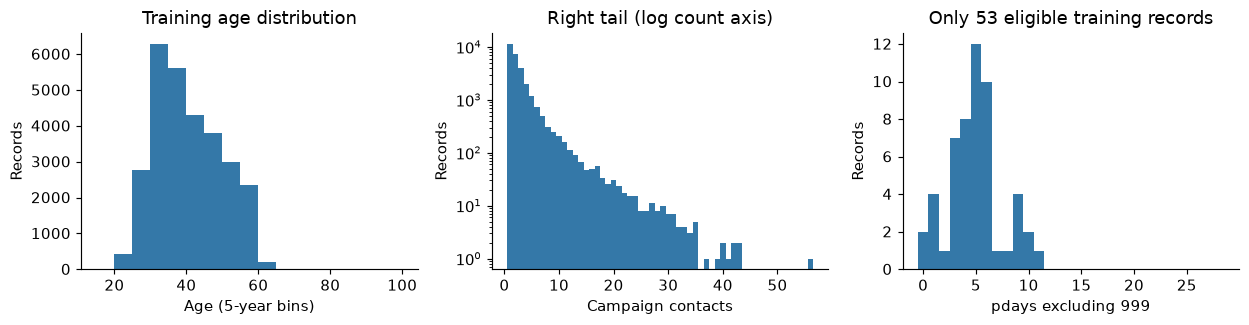

In [3]:
outliers = []
for field in ['age', 'campaign', 'previous', 'pdays', 'euribor3m']:
    x = train.loc[train.pdays.ne(999), field] if field == 'pdays' else train[field]
    q1, q3 = x.quantile([.25, .75]); lo, hi = q1-1.5*(q3-q1), q3+1.5*(q3-q1)
    marked = (x < lo) | (x > hi)
    outliers.append([field, len(x), x.skew(), lo, hi, int(marked.sum()),
                     train.loc[x.index[marked], 'y'].eq('yes').mean()])
show(pd.DataFrame(outliers, columns=['field', 'eligible n', 'skewness', 'IQR low',
    'IQR high', 'flagged n', 'flagged yes rate']))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].hist(train.age, bins=np.arange(15, 105, 5), color=COLORS['train'])
axes[0].set(xlabel='Age (5-year bins)', ylabel='Records', title='Training age distribution')
axes[1].hist(train.campaign, bins=np.arange(.5, train.campaign.max()+1.5), color=COLORS['train'])
axes[1].set(xlabel='Campaign contacts', ylabel='Records', yscale='log', title='Right tail (log count axis)')
axes[2].hist(train.loc[train.pdays.ne(999), 'pdays'], bins=np.arange(-.5, 29.5), color=COLORS['train'])
axes[2].set(xlabel='pdays excluding 999', ylabel='Records', title='Only 53 eligible training records')
finish(fig, '01_distributions')

#### IQR boxplots / 数值字段的箱线图

下图只用**train的28,831条记录**，覆盖9个数值预测字段；采用纵向箱体（数值在纵轴），每个面板单独使用原始尺度，未取log、标准化或截尾。类别字段用前后章节的频数／比例图分析，不强行编码后画箱线图；`duration`不进入拨号前预测字段图。

- **箱体**：Q1（25%分位数）至Q3（75%分位数），中间深色线是中位数；IQR＝Q3−Q1。
- **红色水平虚线**：理论篱笆Q1−1.5×IQR、Q3＋1.5×IQR。**须线**止于篱笆内最远的实际观测值，通常不与理论篱笆重合。
- **空心点**：篱笆外的观测；相同取值会重叠，因此同时标注人数和比例，不能按可见点数数记录。它们是待解释的统计标记，不是自动删除对象。
- `pdays`只画53条非999有效间隔，999的排除只发生在该面板的统计计算，不删除数据集记录。`previous`的Q1＝中位数＝Q3＝0，箱体退化为0处的水平线，所有正值被标记，这不是绘图错误。

代码可随Notebook重跑；下方已保存实际运行生成的图。不同字段单位不同，不按箱体的屏幕高度比较重要性；横向箱宽固定，仅用于展示。

C:\Users\forcifer\AppData\Local\Temp\ipykernel_35500\1478056155.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values.to_numpy(), vert=True, widths=.55, whis=1.5,
C:\Users\forcifer\AppData\Local\Temp\ipykernel_35500\1478056155.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values.to_numpy(), vert=True, widths=.55, whis=1.5,
C:\Users\forcifer\AppData\Local\Temp\ipykernel_35500\1478056155.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values.to_numpy(), vert=True, widths=.55, whis=1.5,
C:\Users\forcifer\AppData\Local\Temp\ipykernel_35500\1478056155.py:28: MatplotlibDeprecationWarning: vert: bool was depre

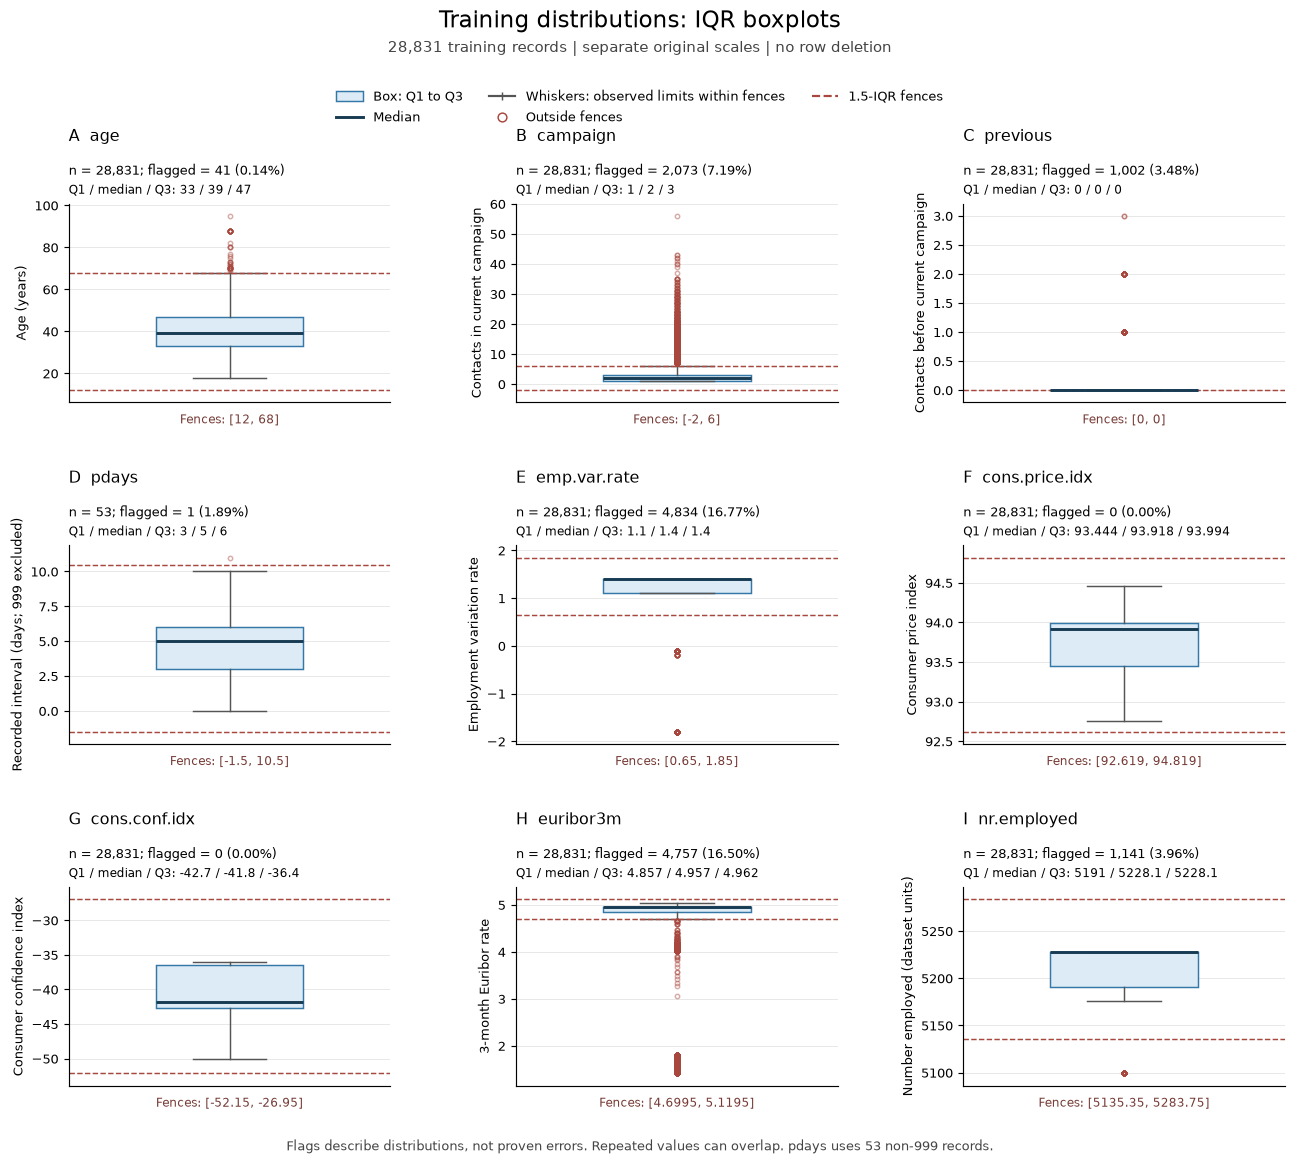

In [ ]:
# Training-only, original-scale boxplots. Fences are NOT deletion rules.
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

iqr_fields = [
    ('age', 'Age (years)'),
    ('campaign', 'Contacts in current campaign'),
    ('previous', 'Contacts before current campaign'),
    ('pdays', 'Recorded interval (days; 999 excluded)'),
    ('emp.var.rate', 'Employment variation rate'),
    ('cons.price.idx', 'Consumer price index'),
    ('cons.conf.idx', 'Consumer confidence index'),
    ('euribor3m', '3-month Euribor rate'),
    ('nr.employed', 'Number employed (dataset units)'),
]
iqr_boxplot_stats = []
fig, axes = plt.subplots(3, 3, figsize=(12.8, 11.2))
for panel, (ax, (field, label)) in enumerate(zip(axes.flat, iqr_fields)):
    # Exclude the sentinel only in this panel; do not remove any dataset rows.
    values = train.loc[train.pdays.ne(999), field] if field == 'pdays' else train[field]
    q1, median, q3 = values.quantile([.25, .5, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = (values < lower) | (values > upper)
    iqr_boxplot_stats.append({
        'field': field, 'n': len(values), 'q1': q1, 'median': median, 'q3': q3,
        'iqr': iqr, 'lower': lower, 'upper': upper, 'flagged': int(flagged.sum())})
    ax.boxplot(values.to_numpy(), vert=True, widths=.55, whis=1.5,
               autorange=False, showfliers=True, patch_artist=True,
               boxprops={'facecolor': '#DCEBF5', 'edgecolor': '#3478A8'},
               medianprops={'color': '#173B53', 'linewidth': 2},
               whiskerprops={'color': '#555555'}, capprops={'color': '#555555'},
               flierprops={'marker': 'o', 'markersize': 3, 'markerfacecolor': 'none',
                           'markeredgecolor': '#A8473D', 'alpha': .45})
    for fence in dict.fromkeys([lower, upper]):
        ax.axhline(fence, color='#A8473D', ls='--', lw=1)
    bottom, top = min(values.min(), lower), max(values.max(), upper)
    padding = .07 * (top-bottom) if top > bottom else 1
    ax.set_ylim(bottom-padding, top+padding)
    ax.set_xlim(.4, 1.6)
    ax.set_xticks([])
    ax.ticklabel_format(axis='y', style='plain', useOffset=False)
    ax.tick_params(axis='y', labelsize=9)
    ax.set_title(f'{chr(65+panel)}  {field}', loc='left', fontsize=11, pad=43)
    ax.set_ylabel(label, fontsize=9)
    ax.text(0, 1.13, f'n = {len(values):,}; flagged = {flagged.sum():,} '
            f'({100*flagged.mean():.2f}%)', transform=ax.transAxes, va='bottom', fontsize=9)
    ax.text(0, 1.035, f'Q1 / median / Q3: {q1:g} / {median:g} / {q3:g}',
            transform=ax.transAxes, va='bottom', fontsize=8.5)
    ax.set_xlabel(f'Fences: [{lower:.6g}, {upper:.6g}]', fontsize=8.5, color='#753A35', labelpad=8)
    ax.set_axisbelow(True)
    ax.grid(axis='y', color='#DADADA', lw=.6, alpha=.7)

fig.suptitle('Training distributions: IQR boxplots', fontsize=16, y=.985)
fig.text(.5, .949, '28,831 training records | separate original scales | no row deletion',
         ha='center', fontsize=10, color='#444444')
fig.legend(handles=[
    Patch(facecolor='#DCEBF5', edgecolor='#3478A8', label='Box: Q1 to Q3'),
    Line2D([], [], color='#173B53', lw=2, label='Median'),
    Line2D([], [], color='#555555', marker='|', label='Whiskers: observed limits within fences'),
    Line2D([], [], marker='o', markerfacecolor='none', color='#A8473D', ls='none', label='Outside fences'),
    Line2D([], [], color='#A8473D', ls='--', label='1.5-IQR fences'),
], loc='upper center', bbox_to_anchor=(.5, .927), ncol=3, frameon=False, fontsize=9)
fig.subplots_adjust(left=.075, right=.98, bottom=.07, top=.82, hspace=.72, wspace=.39)
fig.text(.5, .015, 'Flags describe distributions, not proven errors. Repeated values can overlap. '
         'pdays uses 53 non-999 records.', ha='center', fontsize=9, color='#444444')
# Preserve custom spacing; finish() would replace it with tight_layout().
FIGURES.append(('01b_iqr_boxplots', fig))
plt.show()
plt.close(fig)


**从异常标记到处理决策。** 下表恢复原检查的关键依据；人数均为固定train中的描述统计，不能解释为删行后的模型效果。

| 字段／标记 | 观察到什么 | 为什么保留；应注意什么 |
|---|---|---|
| `age > 68` | 41条，其中38条职业为retired、18条yes（43.90%） | 高龄与退休在语义上相容，尚无录入错误证据；机械删除会排除这部分真实可能存在的人群。样本很少，不能把43.90%当稳定转化率 |
| `campaign > 6` | 2,073条，其中84条yes（4.05%）；计数右长尾 | 较多联系是可解释的业务状态，观察到的低订购率不等于数据无效，也不证明联系导致拒绝；后续联系版使用 `log1p` 表达递减变化 |
| `previous > 0` | Q1=Q3=0，IQR=0；所有1,002条非零历史记录均被标记 | 这是零膨胀计数导致的规则退化；直接删除将丢掉全部有历史联系的记录。后续使用0/1/2+分组，并保留 `poutcome` |
| `pdays` 的有效天数 | 非999仅53条，按有效值计算IQR只标记1条 | 若把999也纳入，篱笆会退化为[999,999]，反而把全部有效天数标成异常。999是特殊编码，不能当999天或普通缺失数值自动填补；具体表示见第3、4节 |
| 宏观指标 | `euribor3m` 标记4,757条；`emp.var.rate` 和 `nr.employed` 分别4,834、1,141条 | 同一时期的宏观值由许多记录共享，标记可能来自经济阶段和窄IQR；不能因此把整个经济阶段当作错误删掉 |

**保留依据是缺乏足够的错误证据，不是“该组yes较多就保留”。** 对yes和no执行相同规则。标记组的订购率用于描述可能失去的覆盖，不作为按标签选择删行的标准。后续审计还发现，按train篱笆，val的上述三个宏观字段均会把整段6,178条记录标记出来；这支持检查时期变化，而非删除验证记录。IQR外、训练值域外、业务上不可能，是三种不同判断。

### 2.4 Skewness and limits / 偏态为什么不等于必须纠正

逻辑回归不要求每个输入服从正态分布。`StandardScaler` 只改变中心和尺度，不消除偏度；非负右偏计数可通过 `log1p` 或平方根压缩长尾，平方／立方通常会放大右尾。是否采用变换要看关系表示、拟合稳定性和验证表现，不能以“看起来更像正态”验收。宏观指标的负偏也不能成为直接取log或开平方的理由，尤其不能忽略负值及字段含义。

最初A/B保留计数原形（B再标准化）；后续联系版才引入 `campaign_log`、`previous`分组、年龄样条等表示。因此，不应把后期特征工程写成最初已经采取的清洗。当前没有按异常标记删行或截尾后重训的对照，也未完成逐条高影响记录、数据来源真实性及客户身份核实；**“暂保留并说明边界”不等于“异常检查已经穷尽”或“删除一定变差”。**

## 3. Focused EDA / 有证据的非显然发现
### 3.1 Shared missingness can inflate association / 共同缺失改变关联

housing和loan的unknown出现在同一批记录中。下面同时计算全部类别和双已知子集的Cramér’s V，
并列出各自分母。剔除unknown会改变人群和类别维度；后一个V不能称为“校正后的真实总体关联”。

In [4]:
from scipy.stats import chi2_contingency
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    denominator = ct.to_numpy().sum() * min(ct.shape[0]-1, ct.shape[1]-1)
    return np.sqrt(chi2_contingency(ct, correction=False)[0]/denominator) if denominator else np.nan
assert train.housing.eq('unknown').equals(train.loan.eq('unknown'))
known = train.housing.ne('unknown') & train.loan.ne('unknown')
association = pd.DataFrame([
    ['housing × loan: all', len(train), cramers_v(train.housing, train.loan)],
    ['housing × loan: both known', int(known.sum()), cramers_v(train.loc[known,'housing'], train.loc[known,'loan'])]],
    columns=['comparison', 'n', 'Cramers V'])
show(association)
show(pd.crosstab(train.poutcome, train.pdays.eq(999)).rename(columns={False:'pdays != 999', True:'pdays = 999'}).reset_index())
print('previous=0 and poutcome=nonexistent agree:',
      bool(train.previous.eq(0).equals(train.poutcome.eq('nonexistent'))))

comparison,n,Cramers V
housing × loan: all,28831,0.7079
housing × loan: both known,28137,0.0486


poutcome,pdays != 999,pdays = 999
failure,3,949
nonexistent,0,27829
success,50,0


previous=0 and poutcome=nonexistent agree: True


**历史字段不能机械互换。** 字典将 `pdays=999` 解释为此前未联系的特殊取值，但本train中，`previous=0` 与 `poutcome=nonexistent` 重合27,829条；`failure` 中却有949条999和3条非999，`success`的50条均非999。这些交叉关系说明，不能直接把三个字段当成完全相同的历史定义。

记录范围、缺失间隔或采集处理差异都可能解释这种现象，目前无法确定机制。因此衍生变量采用“pdays是否999／是否有非999间隔”的中性命名，不将 `pdays_known` 解释为“客户全部历史已知”，也不把999擅自改成一个估计的真实间隔。第4节区分A保留原值、B初版删除与B_pdays拆分；三者是候选表示，不能把删字段当作已经证实没有价值。

### 3.2 Rates, denominators and coverage / 比例、人数与覆盖

组内订购率回答“该组多容易订购”，组人数回答“规模多大”，yes覆盖回答“全部订购者中有多少来自该组”。
总体比例已经是各组比例按人数加权的均值，无须再对组内比例乘一次占比。
下图train/val各用自己的基线；小样本只作为线索，不能由高比例直接指定模型权重。

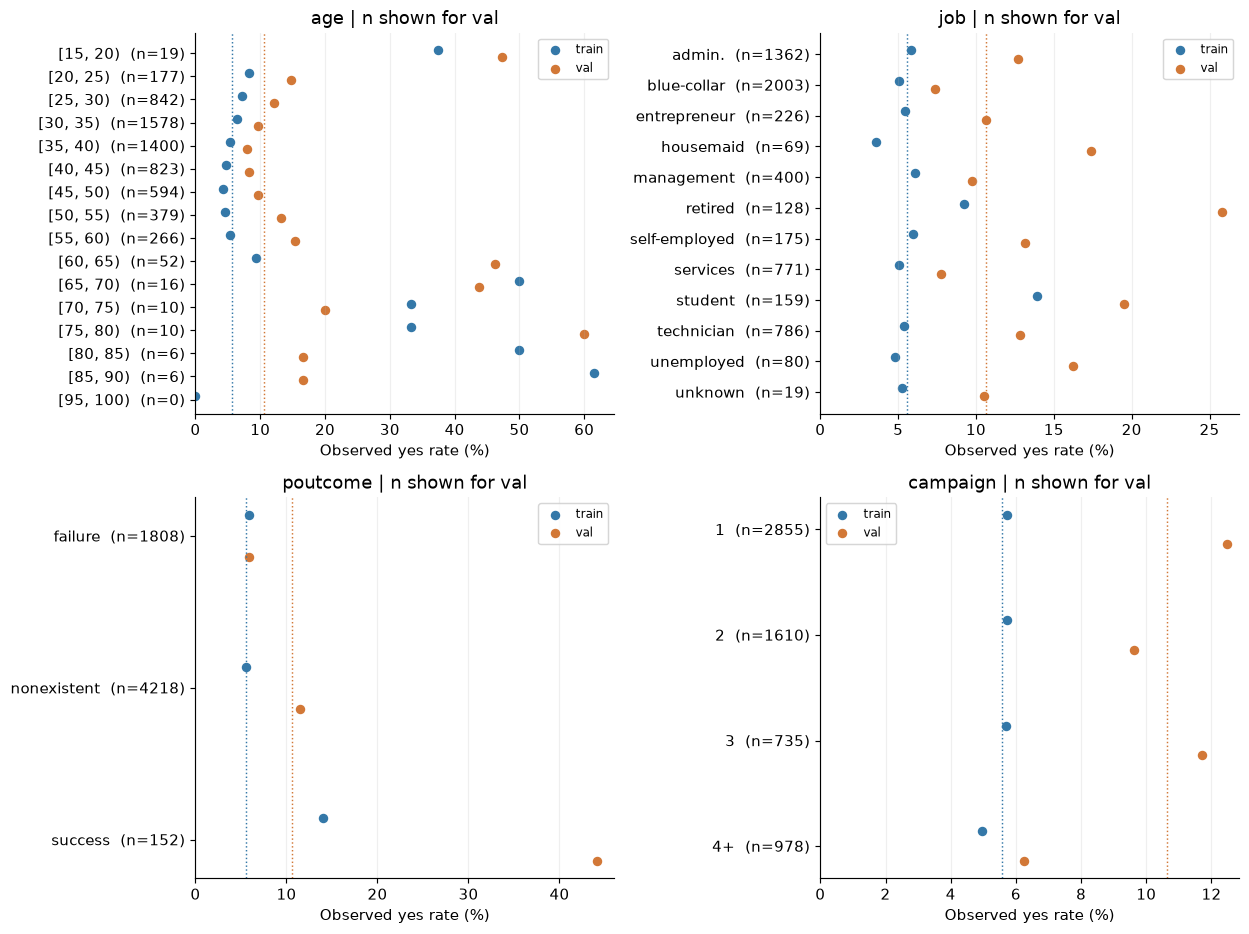

level,n,yes,rate,population share,yes coverage
failure,1808,106,0.0586,0.2927,0.1611
nonexistent,4218,485,0.1150,0.6827,0.7371
success,152,67,0.4408,0.0246,0.1018


In [5]:
def group_label(frame, field):
    if field == 'age': return pd.cut(frame.age, bins=np.arange(15, 105, 5), right=False).astype(str)
    if field == 'campaign': return frame.campaign.map(lambda x: str(x) if x < 4 else '4+')
    return frame[field].astype(str)
def grouped(frame, field):
    g = pd.DataFrame({'level': group_label(frame, field), 'yes': frame.y.eq('yes').astype(int)})
    out = g.groupby('level', sort=True).yes.agg(['size','sum','mean'])
    out.columns = ['n','yes','rate']
    out['population share'] = out.n/len(frame)
    out['yes coverage'] = out.yes/out.yes.sum()
    assert np.isclose((out.rate*out['population share']).sum(), frame.y.eq('yes').mean())
    return out
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, field in zip(axes.flat, ['age','job','poutcome','campaign']):
    gt, gv = grouped(train,field), grouped(val,field)
    levels = list(dict.fromkeys(gt.index.tolist()+gv.index.tolist()))
    if field == 'age': levels = sorted(levels, key=lambda s: int(s.split(',')[0][1:]))
    pos = np.arange(len(levels))
    for delta, label, tab in [(-.14,'train',gt),(.14,'val',gv)]:
        tmp = tab.reindex(levels)
        ax.scatter(tmp.rate*100, pos+delta, label=label, color=COLORS[label], s=30)
        ax.axvline((y_train if label=='train' else y_val).mean()*100, color=COLORS[label], ls=':', lw=1)
    labels=[f'{level}  (n={int(gv.loc[level,"n"]) if level in gv.index else 0})' for level in levels]
    ax.set(yticks=pos, yticklabels=labels, xlabel='Observed yes rate (%)', title=field+' | n shown for val')
    ax.invert_yaxis(); ax.set_xlim(left=0); ax.grid(axis='x', alpha=.2)
    ax.legend(fontsize=8, loc='best')
finish(fig, '02_group_rates')
show(grouped(val, 'poutcome').reset_index())

学生、退休及部分青年/高龄组的比例较高，但不是同一群体，不能把重叠特征当独立证据相加。
val历史success组订购率44.08%，却仅覆盖全部yes的10.18%；nonexistent组比例11.50%，覆盖73.71%。
只关注“最容易买”的小群体会限制召回。campaign的4+组两段均较低，但1/2/3并非严格单调，
只能说“联系次数较多者观察到较低订购率”，不能说多联系导致拒绝。

housing/loan单变量差异较小；default的no/unknown有差异，真实yes样本极少。
month和weekday与阶段、客户选择混在一起：train星期峰值与val不同，不能推荐某个星期打电话来保证效果。

### 3.3 Macro structure and shift / 宏观结构与跨期变化

CPI是价格指数水平，不是通胀率；CCI是消费者信心指标，不是概率。数据字典未给出基期、精确系列代码及发布时点。
train中CPI与CCI **线性相关性弱**（Pearson r≈0.0577），但不能推出统计独立或二者均无预测作用。
其他宏观列存在多重共线性；L2可稳定参数，却不消除相关或保证未来有效。

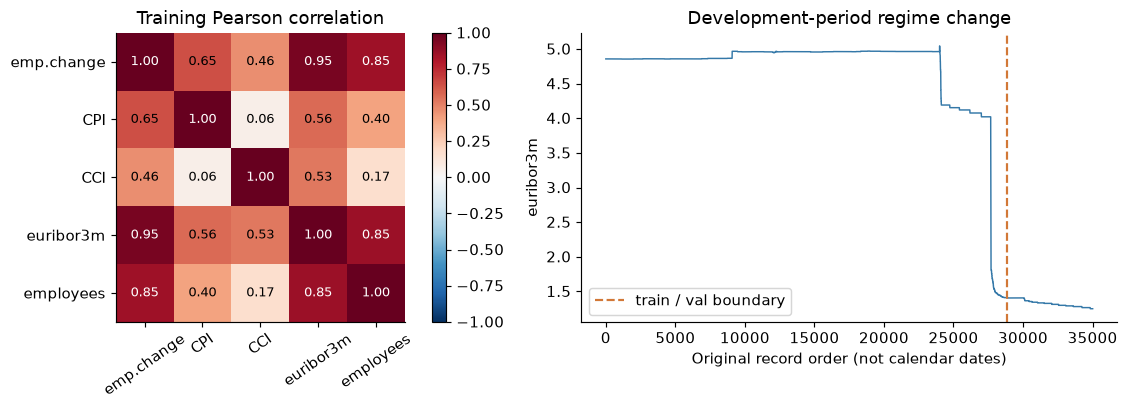

CPI–CCI Pearson r: 0.0576927123923388
Validation euribor outside train range: 6129 / 6178


In [6]:
MACRO = ['emp.var.rate','cons.price.idx','cons.conf.idx','euribor3m','nr.employed']
corr = train[MACRO].corr()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
im=axes[0].imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
short=['emp.change','CPI','CCI','euribor3m','employees']
axes[0].set(xticks=range(5), xticklabels=short, yticks=range(5), yticklabels=short, title='Training Pearson correlation')
axes[0].tick_params(axis='x', rotation=35)
for i in range(5):
    for j in range(5): axes[0].text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=9,color='white' if abs(corr.iloc[i,j])>.7 else 'black')
fig.colorbar(im, ax=axes[0], fraction=.045)
axes[1].plot(dev.index, dev.euribor3m, lw=1, color='#3478A8')
axes[1].axvline(28831, color='#D27837', ls='--', label='train / val boundary')
axes[1].set(xlabel='Original record order (not calendar dates)', ylabel='euribor3m', title='Development-period regime change')
axes[1].legend()
finish(fig, '03_macro_structure')
print('CPI–CCI Pearson r:', corr.loc['cons.price.idx','cons.conf.idx'])
print('Validation euribor outside train range:',
      (~val.euribor3m.between(train.euribor3m.min(),train.euribor3m.max())).sum(), '/', len(val))

## 4. Preparation decisions and mappings / 编码与处理决策

下表保留最初A/B设计，不因后续结果倒改理由。两个方案均排除duration，使用同一种L2逻辑回归。
B同时改变多项，只能解释总处理效果；其后单因素恢复对照负责拆解。

| 项目 | A：最少处理 | B：系统处理初版 | 理由、损失及对照 |
|---|---|---|---|
| 类别 | 完整one-hot，unknown保留 | 一般类别同A | 不给名义类别任意大小顺序 |
| 数值 | 原值 | train标准化 | 影响L2的有效惩罚；A_scaled单独检验缩放 |
| housing/loan | 分别完整one-hot | 两个yes指示+共享unknown | 必须验证两列unknown同步；不是unknown→no |
| default | no/yes/unknown | 仅unknown指示 | yes与no合并，有信息损失；B_default3恢复三类 |
| pdays | 原值含999 | 删除 | train有效记录53条；B_pdays恢复哨兵+中心化有效天数 |
| month | 保留 | 删除 | 季节与时期难分离；B_month恢复 |
| 宏观 | 五列全部保留 | CPI、CCI、euribor3m | 共线性驱动候选删减；B_macro_all恢复五列 |
| 重复/异常 | 保留 | 保留 | 未确认数据错误，不自动删除 |
| 不平衡 | 不加权 | 不加权 | 先固定基线；之后进行独立配对实验 |

**映射示例。** `(housing,loan)=(no,no)/(yes,no)/(no,yes)/(yes,yes)/(unknown,unknown)`
分别映射为`(0,0,0)/(1,0,0)/(0,1,0)/(1,1,0)/(0,0,1)`。
任一列单独unknown时报错。`default_unknown=0`表示“已知”，不是“无违约”。
B_pdays使用`is999`与`d−m_train`；999位置天数置0，指标保留差异；train无有效天数则禁用天数列。
未见类别预设为全零one-hot，不从val学习新词表。

### 4.1 Why these candidates? / 候选处理的依据与信息损失

| 决策 | 当时的依据 | 必须保留的限制 |
|---|---|---|
| B合并 `default` 的yes/no | train中真实yes仅3条，绝大多数为no或unknown，故设计“已知／未知”简化候选 | 这会丢失真实违约状态，不能说yes不可学习或没有意义；val没有yes，`B_default3`也不能验证对该罕见类别的迁移效果 |
| B初版删 `pdays`，并另设拆分对照 | train仅53条非999（约0.18%），有效间隔参数可能不稳定 | 稀少不是无信息证明。A仍把999作为数值保留，是最少处理比较基线，不能将其解释成真实999天 |
| `B_pdays` 使用指示＋中心化天数 | 有效天数减train中位数5，999位置置0且另有 `is999=1` | 置0只是设计矩阵占位，不是认定真实间隔为0。有效天数保留天数单位，不再对大量占位0一起标准化；后来联系版的log表示是另一个方案 |
| B删 `month`、删两列宏观指标 | train内月名与活动阶段难区分，宏观列又存在多重共线性，故提出简化候选 | 不证明月份或宏观信息无用；分别用 `B_month`、`B_macro_all` 恢复。L2缩小系数，但不自动删列、不消除相关，更不保证因果解释 |
| 保留稀有类别及名义类别one-hot | 学生、退休、文盲等都有独立语义；样本少或单变量差异弱不自动成为删类理由 | 不按组内订购率手工给学生／退休“加权”。系数由联合模型拟合；重叠背景和小样本会限制解释，完整one-hot的类别比较使用系数差 |

`housing/loan`的联合编码只在“unknown逐行同步”成立时保留该状态信息；遇到一列未知、一列已知时显式报错。该检查不代表未来永远符合此前提。`B_pdays`中999与中位数5都会出现天数列0，但指示列不同，因此可区分；若训练没有有效间隔，则禁用天数列，而非从val/test估计中心。

### 4.2 Decision rule / 不靠显著性阈值怎样做决策

先由**语义与预测时点**排除不可用信息（如 `duration`），再由train的覆盖、分布、冗余和复杂度提出少量候选。Cramér’s V、相关系数和VIF用于描述及提出假设，不按p值或单一阈值自动删字段；“线性相关性弱”也不是“没有任何关系”。同一模型的单因素恢复／删减才用于讨论某项处理的预测影响；A与B同时改了多项，不能将总差异归给其中一项。

原核心轮次在train拟合、val按预定ROC-AUC/AP等口径选方案及阈值，冻结后报告test；后续已看过原test的探索在第7节另行披露。比较填补、编码、缩放或采样时，数据驱动参数及采样均限于相应训练窗，保留val/test的自然构成，不通过删掉难预测记录或平衡评价集来改善成绩。初版不加权用于固定基线，后续不平衡实验见第9节。

## 5. Core experiment: same logistic model / 同模型比较

$$p_i=\sigma(\beta_0+\phi(x_i)^T\beta),\qquad
L=\sum_i[-y_i\log p_i-(1-y_i)\log(1-p_i)]+\frac{\|\beta\|_2^2}{2C}.$$

$\phi$是各方案的编码；原始变量允许经确定性转换，线性作用发生在变换后的logit空间。
本节C=1、lbfgs、tol=1e-4、L2、无类别权重、截距不惩罚；全部候选统一迭代上限，
若任一达到5000上限则全部以20000重试。截距不简单等于训练基础率的logit。

原规则以val ROC-AUC优先、AP次之、维度/名称破平局；原选择为A_scaled。
所有候选统一报告0.5及val最大F1阈值，F1平局取高阈值。
阈值只改变判类，不改变AUC/AP；同一val优化出的F1含选择乐观性。

下方代码保留完整映射与Pipeline；唯一数据驱动拟合均发生在train。

### 5.1 七个模型究竟哪里不同？

下面都是同一种L2逻辑回归，差别主要在输入表示。`features` 是**预处理后的设计矩阵列数**，不包含截距，不是原始字段数或重要因素个数。

| Model | 相对基线的建模变化 | 本次train编码后features |
|---|---|---:|
| A | 19个原始输入字段；10个类别列完整one-hot，9个数值列原尺度 | 61 |
| A_scaled | 相对A，仅把9个数值列用train均值/标准差缩放 | 61 |
| B | 以4节方案处理unknown；删除month和pdays；宏观只留CPI/CCI/euribor；数值缩放 | 44 |
| B_macro_all | 相对B，恢复emp.var.rate和nr.employed两列 | 46 |
| B_month | 相对B，恢复month；train中9个水平扩展成9列 | 53 |
| B_pdays | 相对B，增加pdays是否999和有效天数中心化两列 | 46 |
| B_default3 | 相对B，将1列default_unknown恢复为default的3列one-hot | 46 |

例如，A的10个类别字段变成52列，加9个数值列得到61；B是34个类别哑变量＋6个连续列＋4个二元列＝44。
`A_scaled` 只改变数值尺度，因此列数不变；删字段、合并编码、恢复类别或把年龄换成多列样条都会改变列数。
不同时间窗若见到的类别不同，列数也可能不同。类别和样条结点仅从各自train学习，不能用val/test补齐类别。

**公平性解释：** 同C固定了超参数，但缩放、维度和特征相关性会改变L2的有效约束，不代表各表示受到完全相同的惩罚。更多features也不等于更强的预测能力。


In [7]:
"""Bank Marketing: explicit feature mappings and reproducible train/validation experiments.
No training or test evaluation occurs at import. Notebook Section 7 owns the protocol.
"""
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss,
    brier_score_loss, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
    precision_recall_curve)
from sklearn.exceptions import ConvergenceWarning
from scipy.special import expit
from threadpoolctl import threadpool_limits

# 编码与显式列组：不拟合分类器；所有数据驱动参数只能来自train。
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

A_CATEGORICAL = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome"]
A_NUMERIC = ["age", "campaign", "pdays", "previous", "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
B_CATEGORICAL = ["job", "marital", "education", "contact", "day_of_week", "poutcome"]
B_CONTINUOUS = ["age", "campaign", "previous", "cons.price.idx", "cons.conf.idx", "euribor3m"]
B_BINARY = ["housing_yes", "loan_yes", "housing_loan_unknown", "default_unknown"]

def encode_target(y):
    if not y.isin(["yes", "no"]).all():
        raise ValueError("Target must contain only yes/no")
    return y.map({"no": 0, "yes": 1}).astype("int8").rename("y_binary")

def valid_pdays(d):
    days = pd.to_numeric(d["pdays"], errors="raise")
    if not np.isfinite(days.to_numpy(dtype=float)).all() or (days < 0).any():
        raise ValueError("pdays must be finite and nonnegative; 999 is the sentinel")
    return days

def learn_pdays_center(train_data):
    days = valid_pdays(train_data)
    valid = days[days.ne(999)]
    return {"center": float(valid.median()) if len(valid) else 0.0,
            "days_enabled": bool(len(valid)), "valid_count": int(len(valid)),
            "scaling": "none_after_train_median_centering"}

def encode_pdays(d, train_non999_median, days_enabled=True):
    if not np.isscalar(train_non999_median):
        raise ValueError("pdays center must be a finite scalar")
    try:
        center = float(train_non999_median)
    except (TypeError, ValueError):
        raise ValueError("pdays center must be a finite scalar") from None
    if not np.isfinite(center):
        raise ValueError("pdays center must be finite")
    days = valid_pdays(d)
    is999 = days.eq(999)
    centered = (days - center).where(~is999, 0.0)
    if not days_enabled:
        centered = pd.Series(0.0, index=d.index)
    return pd.DataFrame({"pdays_is_999": is999.astype("int8"),
                         "pdays_days_centered": centered}, index=d.index)

def prepare_b_features(d, pdays_mode="drop", pdays_center=None, days_enabled=True,
                       keep_month=False, macro_all=False, default_three=False):
    """B默认方案及明确的单因素开关；保持行索引，不修改输入，不使用y。"""
    if pdays_mode not in {"drop", "split"}:
        raise ValueError("pdays_mode must be drop or split")
    x = d.drop(columns=["y", "duration"], errors="ignore").copy()
    for col in ["housing", "loan", "default"]:
        if not x[col].isin(["yes", "no", "unknown"]).all():
            raise ValueError(f"Unexpected category in {col}")
    hu, lu = x["housing"].eq("unknown"), x["loan"].eq("unknown")
    if not hu.equals(lu):
        raise ValueError("housing/loan unknown mismatch: revise encoding explicitly")
    x["housing_yes"] = x["housing"].eq("yes").astype("int8")
    x["loan_yes"] = x["loan"].eq("yes").astype("int8")
    x["housing_loan_unknown"] = hu.astype("int8")
    drop = ["housing", "loan", "pdays"]
    if not default_three:
        x["default_unknown"] = x["default"].eq("unknown").astype("int8")
        drop.append("default")
    if not keep_month:
        drop.append("month")
    if not macro_all:
        drop.extend(["emp.var.rate", "nr.employed"])
    if pdays_mode == "split":
        x = x.join(encode_pdays(d, pdays_center, days_enabled))
    return x.drop(columns=drop)

def make_preprocessor(arm="B", pdays_mode="drop", keep_month=False, macro_all=False, default_three=False):
    """仅构造预处理器；fit时只传train。显式分组，不依赖dtype。"""
    if arm == "A":
        if pdays_mode != "drop" or keep_month or macro_all or default_three:
            raise ValueError("A uses original columns; B-only flags are invalid")
        return ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore", drop=None), A_CATEGORICAL),
            ("num", "passthrough", A_NUMERIC)], remainder="drop")
    if arm != "B" or pdays_mode not in {"drop", "split"}:
        raise ValueError("Invalid arm or pdays_mode")
    categorical = B_CATEGORICAL + (["month"] if keep_month else []) + (["default"] if default_three else [])
    continuous = B_CONTINUOUS + (["emp.var.rate", "nr.employed"] if macro_all else [])
    binary = [c for c in B_BINARY if not (default_three and c == "default_unknown")]
    if pdays_mode == "split":
        binary = binary + ["pdays_is_999"]
    groups = [("cat", OneHotEncoder(handle_unknown="ignore", drop=None), categorical),
              ("num", StandardScaler(), continuous), ("binary", "passthrough", binary)]
    if pdays_mode == "split":
        groups.append(("pdays_days", "passthrough", ["pdays_days_centered"]))
    return ColumnTransformer(groups, remainder="drop")


CANDIDATES = {
    "A": {"arm": "A"},
    "A_scaled": {"arm": "A", "scale_a": True},
    "B": {"arm": "B"},
    "B_macro_all": {"arm": "B", "macro_all": True},
    "B_month": {"arm": "B", "keep_month": True},
    "B_pdays": {"arm": "B", "pdays_mode": "split"},
    "B_default3": {"arm": "B", "default_three": True},
}

class MarketingFeatures(TransformerMixin, BaseEstimator):
    """Train-only data-dependent mapping inside the saved Pipeline."""
    def __init__(self, arm="B", pdays_mode="drop", keep_month=False, macro_all=False, default_three=False):
        self.arm=arm; self.pdays_mode=pdays_mode; self.keep_month=keep_month
        self.macro_all=macro_all; self.default_three=default_three
    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame) or "y" in X or "duration" in X:
            raise ValueError("Pass raw feature DataFrame without target/duration")
        self.feature_names_in_=np.asarray(X.columns,dtype=object)
        self.n_features_in_=X.shape[1]
        self.training_rows_=len(X)
        self.pdays_params_=learn_pdays_center(X) if self.pdays_mode=="split" else None
        self.output_columns_=self._transform(X).columns.tolist()
        return self
    def _transform(self, X):
        if self.arm=="A":
            return X.loc[:,A_CATEGORICAL+A_NUMERIC].copy()
        params=self.pdays_params_ or {"center":None,"days_enabled":True}
        return prepare_b_features(X,pdays_mode=self.pdays_mode,pdays_center=params["center"],
            days_enabled=params["days_enabled"],keep_month=self.keep_month,
            macro_all=self.macro_all,default_three=self.default_three)
    def transform(self, X):
        if not hasattr(self,"output_columns_"):
            raise ValueError("Feature builder is not fitted")
        if "y" in X or "duration" in X:
            raise ValueError("Target/duration must not enter pipeline")
        result=self._transform(X)
        if result.columns.tolist()!=self.output_columns_:
            raise ValueError("Feature order changed")
        return result
    def get_feature_names_out(self,input_features=None):
        return np.asarray(self.output_columns_,dtype=object)

def build_pipeline(spec,max_iter=5000):
    options={k:v for k,v in spec.items() if k!="scale_a"}
    pre=make_preprocessor(**options)
    if spec.get("scale_a",False):
        pre.set_params(transformers=[("cat",OneHotEncoder(handle_unknown="ignore",drop=None),A_CATEGORICAL),
                                    ("num",StandardScaler(),A_NUMERIC)])
    pre.set_params(sparse_threshold=1.0)  # same numerical design, sparse storage for serial CPU fitting
    kwargs=dict(C=1.0,solver="lbfgs",max_iter=max_iter,tol=1e-4,class_weight=None,fit_intercept=True)
    import sklearn
    version=tuple(int(v) for v in sklearn.__version__.split('.')[:2])
    kwargs.update({"l1_ratio":0.0} if version>=(1,8) else {"penalty":"l2"})
    return Pipeline([("features",MarketingFeatures(**options)),("preprocess",pre),
                     ("classifier",LogisticRegression(**kwargs))])

def probabilities(pipe, X):
    classes=pipe.named_steps["classifier"].classes_
    positive=int(np.flatnonzero(classes==1)[0])
    p=pipe.predict_proba(X)[:,positive]
    if not np.isfinite(p).all() or ((p<0)|(p>1)).any():
        raise ValueError("Invalid probabilities")
    return p

def metric_row(y,p,threshold=0.5):
    y=np.asarray(y,dtype=int);p=np.asarray(p,dtype=float)
    if len(y)!=len(p) or not np.isfinite(p).all() or ((p<0)|(p>1)).any():
        raise ValueError("Invalid metric inputs")
    pred=(p>=threshold).astype(int)
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    both=len(np.unique(y))==2
    return {"n":len(y),"positive_rate":float(y.mean()),"mean_probability":float(p.mean()),
      "roc_auc":float(roc_auc_score(y,p)) if both else None,
      "average_precision":float(average_precision_score(y,p)) if both else None,
      "brier":float(brier_score_loss(y,p)),"log_loss":float(log_loss(y,p,labels=[0,1])),
      "threshold":float(threshold),"accuracy":float(accuracy_score(y,pred)),
      "precision":float(tp/(tp+fp)) if tp+fp else np.nan,
      "recall":float(recall_score(y,pred,zero_division=0)),"f1":float(f1_score(y,pred,zero_division=0)),
      "predicted_positive_rate":float(pred.mean()),"tn":int(tn),"fp":int(fp),"fn":int(fn),"tp":int(tp),
      "majority_accuracy_reference":float(max(y.mean(),1-y.mean()))}

def choose_f1_threshold(y,p):
    if len(np.unique(y))!=2:
        raise ValueError("Threshold selection requires both classes in validation")
    precision,recall,thresholds=precision_recall_curve(y,p,drop_intermediate=False)
    score=np.divide(2*precision[:-1]*recall[:-1],precision[:-1]+recall[:-1],
                    out=np.zeros_like(thresholds),where=(precision[:-1]+recall[:-1])>0)
    # Numerical equality tolerance only; not a practical-improvement threshold.
    best=np.flatnonzero(np.isclose(score,score.max(),rtol=0,atol=1e-12))
    return float(thresholds[best[-1]])  # ascending thresholds: prefer higher among tied F1

In [8]:
# All preprocessing and fits use train only. No saved model/results are loaded.
core_models, fit_rows = {}, []
for cap in [5000, 20000]:
    core_models, fit_rows = {}, []
    for name, spec in CANDIDATES.items():
        pipe = build_pipeline(spec, max_iter=cap)
        with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always'); pipe.fit(X_train, y_train)
        it = int(pipe.named_steps['classifier'].n_iter_[0])
        ok = it < cap and not any(issubclass(w.category, ConvergenceWarning) for w in caught)
        core_models[name] = pipe
        fit_rows.append({'model':name,'iterations':it,'converged':ok,
                         'features':len(pipe.named_steps['classifier'].coef_[0])})
    if all(r['converged'] for r in fit_rows): break
assert all(r['converged'] for r in fit_rows), 'Inspect convergence before interpreting results.'
show(pd.DataFrame(fit_rows))
val_prob = {name:probabilities(pipe,X_val) for name,pipe in core_models.items()}
core_rows=[]
for name, pipe in core_models.items():
    for split,xx,yy in [('train',X_train,y_train),('val',X_val,y_val)]:
        core_rows.append({'model':name,'split':split,**metric_row(yy,probabilities(pipe,xx))})
for split,yy in [('train',y_train),('val',y_val)]:
    core_rows.append({'model':'train_prior_dummy','split':split,
                     **metric_row(yy,np.full(len(yy),y_train.mean()))})
core_reference=pd.DataFrame(core_rows)
METRIC_COLUMNS=['model','roc_auc','average_precision','accuracy','precision','recall','f1',
                'log_loss','brier','tp','fp','fn','tn']
show(core_reference[core_reference.split=='val'][METRIC_COLUMNS])


model,iterations,converged,features
A,3853,True,61
A_scaled,36,True,61
B,37,True,44
B_macro_all,34,True,46
B_month,35,True,53
B_pdays,24,True,46
B_default3,27,True,46


model,ROC-AUC,AP,Accuracy,Precision,Recall,F1,Log loss,Brier,tp,fp,fn,tn
A,0.6633,0.2015,0.8935,—,0.0000,0.0000,0.3262,0.0923,0,0,658,5520
A_scaled,0.6650,0.2094,0.8935,—,0.0000,0.0000,0.3226,0.0916,0,0,658,5520
B,0.6206,0.1591,0.8935,—,0.0000,0.0000,0.3546,0.1001,0,0,658,5520
B_macro_all,0.6231,0.1599,0.8935,—,0.0000,0.0000,0.3480,0.0980,0,0,658,5520
B_month,0.6533,0.1919,0.8935,—,0.0000,0.0000,0.3286,0.0928,0,0,658,5520
B_pdays,0.5982,0.1601,0.8907,0.2821,0.0167,0.0316,0.3583,0.1011,11,28,647,5492
B_default3,0.6055,0.1489,0.8935,—,0.0000,0.0000,0.3563,0.1005,0,0,658,5520
train_prior_dummy,0.5000,0.1065,0.8935,—,0.0000,0.0000,0.3588,0.0977,0,0,658,5520


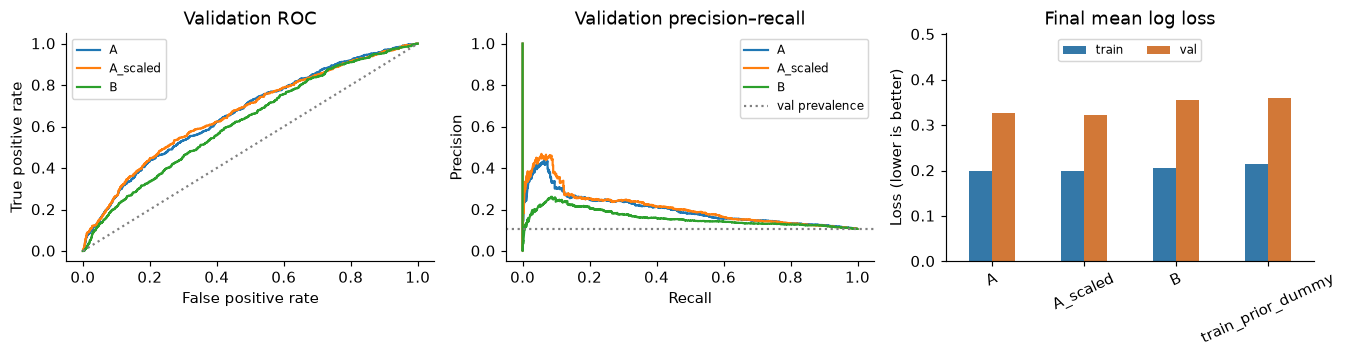

model,rule,threshold,ROC-AUC,AP,Accuracy,Precision,Recall,F1,Log loss,Brier,tp,fp,fn,tn
A,fixed_0.5,0.5000,0.6633,0.2015,0.8935,—,0.0000,0.0000,0.3262,0.0923,0,0,658,5520
A,val_F1_selection_only,0.1510,0.6633,0.2015,0.7601,0.2061,0.4392,0.2806,0.3262,0.0923,289,1113,369,4407
A_scaled,fixed_0.5,0.5000,0.6650,0.2094,0.8935,—,0.0000,0.0000,0.3226,0.0916,0,0,658,5520
A_scaled,val_F1_selection_only,0.1284,0.6650,0.2094,0.7621,0.2104,0.4483,0.2864,0.3226,0.0916,295,1107,363,4413
B,fixed_0.5,0.5000,0.6206,0.1591,0.8935,—,0.0000,0.0000,0.3546,0.1001,0,0,658,5520
B,val_F1_selection_only,0.2161,0.6206,0.1591,0.6727,0.1542,0.4620,0.2312,0.3546,0.1001,304,1668,354,3852
B_macro_all,fixed_0.5,0.5000,0.6231,0.1599,0.8935,—,0.0000,0.0000,0.3480,0.0980,0,0,658,5520
B_macro_all,val_F1_selection_only,0.1919,0.6231,0.1599,0.6186,0.1506,0.5562,0.2370,0.3480,0.0980,366,2064,292,3456
B_month,fixed_0.5,0.5000,0.6533,0.1919,0.8935,—,0.0000,0.0000,0.3286,0.0928,0,0,658,5520
B_month,val_F1_selection_only,0.1526,0.6533,0.1919,0.7569,0.2032,0.4392,0.2779,0.3286,0.0928,289,1133,369,4387


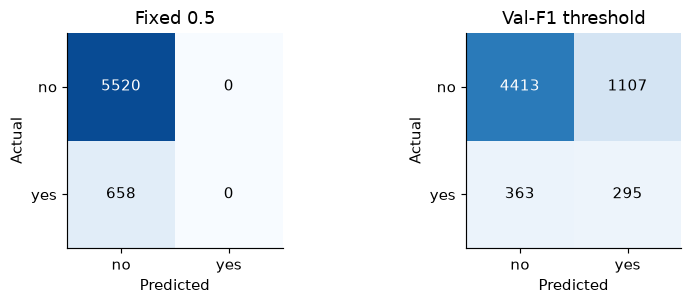

In [9]:
focus = ['A','A_scaled','B']
fig, axes = plt.subplots(1,3,figsize=(13,3.5))
for name in focus:
    p = val_prob[name]
    fpr,tpr,_=roc_curve(y_val,p); axes[0].plot(fpr,tpr,label=name)
    pp,rr,_=precision_recall_curve(y_val,p); axes[1].plot(rr,pp,label=name)
axes[0].plot([0,1],[0,1],':',color='grey')
axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='Validation ROC')
axes[1].axhline(y_val.mean(),ls=':',color='grey',label='val prevalence')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Validation precision–recall')
loss=core_reference[core_reference.model.isin(focus+['train_prior_dummy'])].pivot(index='model',columns='split',values='log_loss').reindex(focus+['train_prior_dummy'])
loss.plot.bar(ax=axes[2],rot=25,color=[COLORS['train'],COLORS['val']])
axes[2].set(title='Final mean log loss',ylabel='Loss (lower is better)',xlabel='',ylim=(0,float(loss.max().max())*1.4))
axes[2].legend(fontsize=8,ncol=2,loc='upper center')
for ax in axes[:2]: ax.legend(fontsize=8)
finish(fig,'04_core_validation')
thresholds={name:choose_f1_threshold(y_val,p) for name,p in val_prob.items()}
selected='A_scaled'
for name in CANDIDATES:
    assert np.isclose(choose_f1_threshold(y_val,val_prob[name]),thresholds[name],atol=1e-12,rtol=0)
val_thresholds=pd.DataFrame([
    {'model':name,'rule':rule,**metric_row(y_val,p,t)}
    for name,p in val_prob.items() for rule,t in [('fixed_0.5',.5),('val_F1_selection_only',thresholds[name])]])
show(val_thresholds[['model','rule','threshold']+METRIC_COLUMNS[1:]])
fig,axes=plt.subplots(1,2,figsize=(8,3))
for ax,t,title in zip(axes,[.5,thresholds[selected]],['Fixed 0.5','Val-F1 threshold']):
    cm=confusion_matrix(y_val,val_prob[selected]>=t,labels=[0,1])
    ax.imshow(cm,cmap='Blues',vmin=0,vmax=len(val));ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['no','yes'],yticklabels=['no','yes'],xlabel='Predicted',ylabel='Actual',title=title)
    for (i,j),value in np.ndenumerate(cm): ax.text(j,i,str(value),ha='center',va='center',color='white' if value>len(val)/2 else 'black')
finish(fig,'05_validation_confusion')

In [10]:
# Full one-hot needs coefficient differences between two levels.
contrast_rows=[]
for name in ['A','A_scaled','B']:
    pipe=core_models[name]
    coef=pd.Series(pipe.named_steps['classifier'].coef_[0],
                   index=pipe.named_steps['preprocess'].get_feature_names_out())
    for reference in ['failure','nonexistent']:
        delta=coef['cat__poutcome_success']-coef['cat__poutcome_'+reference]
        contrast_rows.append({'model':name,'comparison':'success vs '+reference,
                             'conditional_log_odds_difference':delta,'conditional_odds_ratio':np.exp(delta)})
show(pd.DataFrame(contrast_rows))


model,comparison,conditional_log_odds_difference,conditional_odds_ratio
A,success vs failure,0.1673,1.1821
A,success vs nonexistent,-0.1985,0.8199
A_scaled,success vs failure,0.1074,1.1134
A_scaled,success vs nonexistent,0.4446,1.5599
B,success vs failure,1.0815,2.9490
B,success vs nonexistent,0.7675,2.1543


**结果。** A的val AUC/AP为0.6633/0.2015，A_scaled为0.6650/0.2094，B为0.6206/0.1591。
A_scaled的优势很小，不声称稳定胜出；B比A更差，说明合理的清理理由不保证预测收益。
B恢复月份改善最大，但val仅包含apr/may，不能外推为月份在所有时期都有效。
同C控制超参数，不代表不同缩放、维度和参数化的有效正则强度完全等价。

0.5下几乎全判no，Accuracy≈89.35%并不代表找到订购者；A_scaled在val-F1阈值下Recall≈44.83%、Precision≈21.04%。
增加检出伴随误报。损失图显示的是**拟合结束后的train/val平均log loss**，不是逐迭代训练曲线，
两段差异不能只归为过拟合，还可能包含基础率及输入变化。

**系数解释。** 完整one-hot加截距在无惩罚下冗余；L2提供特定参数化下的稳定解。
同一字段类别a对b的条件几率比为exp(βa−βb)，不是exp(βa)。
相关历史字段的条件对比可能缺少实际数据支持；系数、相关性和预测贡献均不是因果效应。

### A/B核心模型原运行：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|A|val|top10|6178|0.1065|—|0.6633|0.2015|0.8423|0.2443|0.2295|0.2367|0.3262|0.0923|151|467|507|5053|
|A_scaled|val|top10|6178|0.1065|—|0.6650|0.2094|0.8423|0.2443|0.2295|0.2367|0.3226|0.0916|151|467|507|5053|
|B|val|top10|6178|0.1065|—|0.6206|0.1591|0.8359|0.2120|0.1991|0.2053|0.3546|0.1001|131|487|527|5033|
|B_macro_all|val|top10|6178|0.1065|—|0.6231|0.1599|0.8343|0.2039|0.1915|0.1975|0.3480|0.0980|126|492|532|5028|
|B_month|val|top10|6178|0.1065|—|0.6533|0.1919|0.8410|0.2379|0.2234|0.2304|0.3286|0.0928|147|471|511|5049|
|B_pdays|val|top10|6178|0.1065|—|0.5982|0.1601|0.8343|0.2039|0.1915|0.1975|0.3583|0.1011|126|492|532|5028|
|B_default3|val|top10|6178|0.1065|—|0.6055|0.1489|0.8310|0.1877|0.1763|0.1818|0.3563|0.1005|116|502|542|5018|
|train_prior_dummy|val|top10|6178|0.1065|—|0.5000|0.1065|0.8109|0.0874|0.0821|0.0846|0.3588|0.0977|54|564|604|4956|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（15行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|A|val|fixed_0.5|6178|0.1065|0.5|0.6633|0.2015|0.8935|—|0.0000|0.0000|0.3262|0.0923|0|0|658|5520|
|A_scaled|val|fixed_0.5|6178|0.1065|0.5|0.6650|0.2094|0.8935|—|0.0000|0.0000|0.3226|0.0916|0|0|658|5520|
|B|val|fixed_0.5|6178|0.1065|0.5|0.6206|0.1591|0.8935|—|0.0000|0.0000|0.3546|0.1001|0|0|658|5520|
|B_macro_all|val|fixed_0.5|6178|0.1065|0.5|0.6231|0.1599|0.8935|—|0.0000|0.0000|0.3480|0.0980|0|0|658|5520|
|B_month|val|fixed_0.5|6178|0.1065|0.5|0.6533|0.1919|0.8935|—|0.0000|0.0000|0.3286|0.0928|0|0|658|5520|
|B_pdays|val|fixed_0.5|6178|0.1065|0.5|0.5982|0.1601|0.8907|0.2821|0.0167|0.0316|0.3583|0.1011|11|28|647|5492|
|B_default3|val|fixed_0.5|6178|0.1065|0.5|0.6055|0.1489|0.8935|—|0.0000|0.0000|0.3563|0.1005|0|0|658|5520|
|train_prior_dummy|val|fixed_0.5|6178|0.1065|0.5|0.5000|0.1065|0.8935|—|0.0000|0.0000|0.3588|0.0977|0|0|658|5520|
|A|val|val_f1|6178|0.1065|0.15103434|0.6633|0.2015|0.7601|0.2061|0.4392|0.2806|0.3262|0.0923|289|1113|369|4407|
|A_scaled|val|val_f1|6178|0.1065|0.1283533|0.6650|0.2094|0.7621|0.2104|0.4483|0.2864|0.3226|0.0916|295|1107|363|4413|
|B|val|val_f1|6178|0.1065|0.21610865|0.6206|0.1591|0.6727|0.1542|0.4620|0.2312|0.3546|0.1001|304|1668|354|3852|
|B_macro_all|val|val_f1|6178|0.1065|0.19193474|0.6231|0.1599|0.6186|0.1506|0.5562|0.2370|0.3480|0.0980|366|2064|292|3456|
|B_month|val|val_f1|6178|0.1065|0.15256322|0.6533|0.1919|0.7569|0.2032|0.4392|0.2779|0.3286|0.0928|289|1133|369|4387|
|B_pdays|val|val_f1|6178|0.1065|0.20304083|0.5982|0.1601|0.5887|0.1397|0.5547|0.2232|0.3583|0.1011|365|2248|293|3272|
|B_default3|val|val_f1|6178|0.1065|0.2023331|0.6055|0.1489|0.5838|0.1411|0.5714|0.2263|0.3563|0.1005|376|2289|282|3231|

</details>


### A/B核心模型原运行：完整性能

下表为每个模型在各前向评价窗的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|A|train|top10|28831|0.0557|—|0.6586|0.1744|0.8756|0.1567|0.2814|0.2013|0.1999|0.0495|452|2432|1154|24793|
|A_scaled|train|top10|28831|0.0557|—|0.6583|0.1740|0.8760|0.1585|0.2846|0.2036|0.1999|0.0495|457|2427|1149|24798|
|B|train|top10|28831|0.0557|—|0.6366|0.1433|0.8714|0.1356|0.2435|0.1742|0.2046|0.0507|391|2493|1215|24732|
|B_macro_all|train|top10|28831|0.0557|—|0.6328|0.1465|0.8724|0.1408|0.2528|0.1808|0.2044|0.0506|406|2478|1200|24747|
|B_month|train|top10|28831|0.0557|—|0.6582|0.1739|0.8756|0.1567|0.2814|0.2013|0.2000|0.0495|452|2432|1154|24793|
|B_pdays|train|top10|28831|0.0557|—|0.6364|0.1428|0.8715|0.1359|0.2441|0.1746|0.2046|0.0507|392|2492|1214|24733|
|B_default3|train|top10|28831|0.0557|—|0.6365|0.1438|0.8715|0.1363|0.2447|0.1751|0.2047|0.0507|393|2491|1213|24734|
|train_prior_dummy|train|top10|28831|0.0557|—|0.5000|0.0557|0.8491|0.0243|0.0436|0.0312|0.2150|0.0526|70|2814|1536|24411|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（8行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|A|train|fixed_0.5|28831|0.0557|0.5|0.6586|0.1744|0.9452|0.6000|0.0486|0.0899|0.1999|0.0495|78|52|1528|27173|
|A_scaled|train|fixed_0.5|28831|0.0557|0.5|0.6583|0.1740|0.9448|0.5620|0.0423|0.0787|0.1999|0.0495|68|53|1538|27172|
|B|train|fixed_0.5|28831|0.0557|0.5|0.6366|0.1433|0.9443|—|0.0000|0.0000|0.2046|0.0507|0|0|1606|27225|
|B_macro_all|train|fixed_0.5|28831|0.0557|0.5|0.6328|0.1465|0.9443|—|0.0000|0.0000|0.2044|0.0506|0|0|1606|27225|
|B_month|train|fixed_0.5|28831|0.0557|0.5|0.6582|0.1739|0.9449|0.5739|0.0411|0.0767|0.2000|0.0495|66|49|1540|27176|
|B_pdays|train|fixed_0.5|28831|0.0557|0.5|0.6364|0.1428|0.9443|1.0000|0.0006|0.0012|0.2046|0.0507|1|0|1605|27225|
|B_default3|train|fixed_0.5|28831|0.0557|0.5|0.6365|0.1438|0.9443|—|0.0000|0.0000|0.2047|0.0507|0|0|1606|27225|
|train_prior_dummy|train|fixed_0.5|28831|0.0557|0.5|0.5000|0.0557|0.9443|—|0.0000|0.0000|0.2150|0.0526|0|0|1606|27225|

</details>


## 6. Test-set evaluation / 测试集评估

本节在预留的测试集上，评估已经冻结的A、B和A_scaled模型。**测试集未参与本轮模型训练、方案选择或阈值确定**；评估直接使用已训练模型和验证集确定的阈值。
A_scaled是验证集选中的方案，A和B作为对照，结果如下。


### A/B核心模型原运行：完整性能

下表为每个模型在test的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|A|test|top10|6179|0.3845|—|0.5632|0.4398|0.6038|0.4417|0.1149|0.1824|0.8366|0.2843|273|345|2103|3458|
|B|test|top10|6179|0.3845|—|0.4690|0.3542|0.5757|0.3010|0.0783|0.1242|0.9728|0.3145|186|432|2190|3371|
|A_scaled|test|top10|6179|0.3845|—|0.5773|0.4466|0.6100|0.4725|0.1229|0.1951|0.8151|0.2752|292|326|2084|3477|
|train_prior_dummy|test|top10|6179|0.3845|—|0.5000|0.3845|0.5358|0.1019|0.0265|0.0421|1.1457|0.3448|63|555|2313|3248|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（7行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|A|test|fixed_0.5|6179|0.3845|0.5|0.5632|0.4398|0.6126|0.4751|0.0724|0.1256|0.8366|0.2843|172|190|2204|3613|
|B|test|fixed_0.5|6179|0.3845|0.5|0.4690|0.3542|0.6155|—|0.0000|0.0000|0.9728|0.3145|0|0|2376|3803|
|A_scaled|test|fixed_0.5|6179|0.3845|0.5|0.5773|0.4466|0.6092|0.4601|0.0947|0.1571|0.8151|0.2752|225|264|2151|3539|
|train_prior_dummy|test|fixed_0.5|6179|0.3845|0.5|0.5000|0.3845|0.6155|—|0.0000|0.0000|1.1457|0.3448|0|0|2376|3803|
|A|test|val_f1|6179|0.3845|0.15103434|0.5632|0.4398|0.5676|0.4454|0.5080|0.4746|0.8366|0.2843|1207|1503|1169|2300|
|B|test|val_f1|6179|0.3845|0.21610865|0.4690|0.3542|0.5661|0.2891|0.0880|0.1349|0.9728|0.3145|209|514|2167|3289|
|A_scaled|test|val_f1|6179|0.3845|0.1283533|0.5773|0.4466|0.5480|0.4435|0.6894|0.5398|0.8151|0.2752|1638|2055|738|1748|

</details>


A_scaled原test AUC≈0.577，跨期区分弱。test正类率约38.45%，全no准确率仍有61.55%。
Precision/AP等随评价人群基础率改变；固定阈值的Recall也可能随条件分布改变，但不能说仅基础率变化就必然改变Recall。
数据支持存在迁移问题，尚不能识别它完全来自标签先验、客户构成还是条件关系变化。

## 7. Post-freeze exploration on test / 冻结测试后的探索：统一 test 展示

**从本节起，所有实验主结果都在同一段 test 上展示；train/val 仅作为拟合、调参和选择依据补充。**
train 为行 `[0,28831)`（28,831人）；val 为 `[28831,35009)`（6,178人）；
test 为 `[35009,41188)`（6,179人，2,376个 yes）。行区间均为0起点、右端不包含。

每条支线使用最终开发阶段已保存的配置与模型，不将D1–D4中间训练检查点当成另一组最终候选。
训练通常只用原train；val用于比较方案、校准或冻结阈值，**没有统一改成 train+val 重训**。
近期窗口模型只用原train末12,000行；早期校准基模型只用原train前80%，各表逐项记录。

**证据性质：POSTHOC_SUPPLEMENTARY_TEST_NOT_INDEPENDENT_CONFIRMATION。**
原test早已被查看，因此这些结果是事后补充评价，不能视为新模型的独立确认。
本次没有在test上fit、搜索参数、选阈值、选窗口或进行标签反馈更新。
Top5/10/20%是预设联系预算；展示排序不等于再次选模。

每节正文最多展示10项；其余候选、0.5/Top5/Top20/已保存开发阈值、分组指标和原开发记录均可展开。
固定阈值无预测正例时Precision记为“—”，F1按zero_division=0；ECE使用10个等宽概率箱。

<details>
<summary>此前的开发轨迹与前向窗口定义（历史记录）</summary>

## 7. Development trajectory / 后续试错为何发生

**以下是第6节测试之后的调整与补测。** 拟合、调参和阈值选择仍限于train/val；但原test结果已经被查看，后续补测属于事后评估，不能再当作新的独立盲测。val也被重复使用，重叠的时间前缀不是独立重复。好结果、无收益和退化都保留，不把后续方案冒充最初预注册方案。

原冻结运行`20261014_200642_059600`先按val选定A_scaled，于2026-10-15完成第6节的A/B/A_scaled测试，沿用原完整精度阈值，没有合并train+val重训。正文的历史结果由已保存预测复算，运行Notebook不会新增test预测。

| 实验阶段 | 为什么做 | 实际对照与结论 | 取舍 |
|---|---|---|---|
| diagnosis | 弱表现来自求解还是信息？ | 检查C、严格tol、log计数、早期年龄样条、近期12000条及时间窗；未有一致大幅提升 | 后续统一严格求解；早期5节点样条不与后期4节点混称 |
| macro | 宏观指标是否主导？ | 全5列/全删/仅3列；val接近，跨窗与事后test不稳定 | 不把宏观判为全部无用 |
| personal_macro | 肉眼发现青年/退休/历史成功较高 | 30候选：年龄表示、联系历史、宏观惩罚、单字段删除 | 职业类别由损失拟合，不手工抬高学生权重 |
| weights | 类别权重与年龄×职业交互能否改善？ | 正类权重1/2/5/balanced及有限交互 | 固定0.5的Recall提升不等于排序提升 |
| early_calibration | 能否修复概率迁移？ | 前80%拟合、后20%校准；缩短训练后历史类别覆盖受损 | 保留失败；与后来的完整train基模型校准分开 |
| scope | 个人背景本身是否足够？ | 七项个人背景 vs 加渠道/联系历史，两者均删日历和宏观 | 联系版更适合已有营销历史的人群 |
| precision | 想提高推荐名单的Precision | 16个LR：两信息范围×两年龄表示×四C；12浅树；Precision目标且人数≥30 | 保存不可达规则；不能只选很少人制造高Precision |
| boosting（附录） | 高分误报是否能被非线性修复？ | 误报群体核查＋8个HGB；没有稳定超过联系LR | 超出课程简单模型主线，不作为主模型 |
| closeout | 结束候选评估并补Accuracy | 111个预测器版本、3参考规则、225行事后测试结果 | 已见test，仅描述，不选test冠军 |
| binning / audit | 检查同学分箱及编码、异常问题 | 8个分箱拟合；早期C=1时pdays分箱AP上升而AUC略降；编码/批次不变性核查 | 不仅凭单一指标替换编码，不删除全部异常 |
| imbalance | 正例过少是否主要瓶颈？ | 395次开发拟合：5个LR各自配对，加3类RF；后授权79模型事后test | 无稳定全面改进，详见9节 |
| calibration | 历史成功概率低，是否应加权/校准？ | 历史列尺度0.5/1/2；4模型×3窗口×2映射×4前向折 | 校准不创造新排序，未加入默认流程 |
| refinement | 最后检查编码、简化、时间权重 | 4版本×5窗共20次拟合；只train/val | 删除贷款项仅小幅收益，其他两项不默认采用 |

**开发窗口的数据范围。** 以下按原始CSV的数据记录顺序，从**第1条记录**开始计数，**不含表头**；“第a–b条”包含两端。编号表示记录位置，不是客户ID或具体日期。

| 窗口 | 用于训练的记录 | 训练记录数 | 用于评价的记录 | 评价记录数 |
|---|---|---:|---|---:|
| D1 | 第1–12,000条 | 12,000条 | 第12,001–16,000条 | 4,000条 |
| D2 | 第1–16,000条 | 16,000条 | 第16,001–20,000条 | 4,000条 |
| D3 | 第1–20,000条 | 20,000条 | 第20,001–24,000条 | 4,000条 |
| D4 | 第1–24,000条 | 24,000条 | 第24,001–28,831条 | 4,831条 |
| val（原验证集） | 第1–28,831条 | 28,831条 | 第28,832–35,009条 | 6,178条 |

例如，D1用前12,000条记录训练，再用紧接着的4,000条记录评价；D2将训练范围扩大到前16,000条，再评价后面的4,000条。这是**训练范围逐渐扩大的前向验证**。D1–D4位于原train范围内，最后的val窗口使用原来的验证段；这些开发窗口均不包含test记录。各窗共享部分训练记录，不能当作彼此独立的重复实验。

**为什么这样划分窗口？** 我们要检查的是“用较早的数据训练，能否预测后面的记录”。因此沿用CSV的记录顺序，每次只用评价段之前的数据训练，训练范围随窗口逐步扩大，模拟历史数据不断积累的情况。这是扩展训练窗口的前向验证，不是每次只保留最近固定条数的滑动窗口；记录顺序用于近似先后关系，不能据此补出具体日期。

只看原val，容易把某一个阶段的好表现当成普遍规律。增加D1–D4，是为了观察同一方案在更早的几个阶段是否也有改善，识别“只在某一段有效”的结果。评价段保留各自真实的正例率和类别构成，不为追求比例一致而重排记录。

**为什么从12,000条开始、每次评价约4,000条？** 这组边界是在起始训练量、评价段大小和实验次数之间的实用取舍：先保留12,000条训练记录，再划出多个后续评价段；D4接收原train剩余的4,831条，最后继续使用原来6,178条的val。这样保留了原70/15/15划分及test边界。12,000和4,000不是理论证明或搜索得到的最优长度，也不代表固定月份或保证各窗正例数、稀有类别覆盖相同。

每窗的编码、缩放等拟合只能使用该窗训练段，再应用到后面的评价段。这种检查能提供跨阶段稳定性的证据，但不能消除已经查看test、反复使用val带来的限制；训练段互相重叠，各窗成绩也不能当作独立重复实验来计算独立重复意义下的置信区间。

各轮已有预测已在本地重新核对指标，下方按阶段保留全部候选。本节按train/val结果比较开发方案；第8.1节另外列出已有的事后测试结果。

**统一读表规则。** ROC-AUC和AP评价概率排序；Brier和log loss评价概率误差；Accuracy、Precision、Recall、F1及混淆计数必须对应选人规则。
下方为所有保存预测补齐`fixed_0.5`与`top10`两种口径，并保留原阈值规则。Top10按分数取前ceil(0.1N)人，同分按原始行号，完全不看标签选人；它是联系预算，不是新的概率阈值优化。
同val选择的F1/Precision阈值标为selection only；previous-window/fit阈值按原来更早的数据确定。历史test只应用已经保存的规则。
`—`表示无人预测为yes时Precision未定义（分母0），或Top10不存在单一含并列处理的概率阈值；不是漏算。

**F1为什么这样计算？** F1是Precision与Recall的**调和平均**，不是普通算术平均。两种常见写法是等价的：

$$P=\mathrm{Precision}=\frac{TP}{TP+FP},\qquad R=\mathrm{Recall}=\frac{TP}{TP+FN},$$

$$F_1=\frac{2PR}{P+R}=\frac{2TP}{2TP+FP+FN}.$$

这里，TP是正确找到的订购者，FP是误报为订购者的人，FN是漏掉的订购者。将上面的P、R代入并约分，就得到右边按人数计算的公式；它仍是同一个F1。F1同时兼顾“找得准”和“找得全”，其中一项很低会拖低得分。TN（正确预测为no）不进入F1，因此大量猜对no不会直接抬高F1；F1也不等于业务收益最优。

若实际存在订购者却全部预测为no，则TP=FP=0、FN>0：Precision未定义而显示`—`，但按人数公式计算F1=0，并不矛盾。若TP=FP=FN=0，则F1本身也未定义，需说明软件约定；本代码采用`zero_division=0`，当前这些含真实正例的评价窗不属于这一情形。

全部比例用0–1表示，不同窗口、样本量和基础率分开报告；不能混成一个总体排名。


</details>


### 7.1 实验覆盖与阅读说明

本次共有 **407 条分节候选引用**，对应 **276 个预测定义**。
同一个模型可能被不同章节重复引用；不能把这些数量当成独立算法数。
复用 193 组历史test概率，只为缺失结果执行
**19 次唯一基模型test预测**；校准输出由冻结参数映射得到。

|实验支线|test配置/参照数|
|---|---|
|求解、正则与早期特征诊断|8|
|严格求解复核|1|
|宏观字段消融|4|
|个人、联系历史与宏观联合设计|31|
|类别权重与年龄×职业交互|16|
|早期时间校准|9|
|信息范围|2|
|LR与浅决策树的Precision约束|30|
|HGB扩展支线|8|
|联系次数／历史分箱|8|
|最后四个单因素方案|4|
|poutcome尺度0.5/1/2|3|
|历史诊断基模型|8|
|五个LR及三类RF不平衡对照|79|
|历史信息校准及常数参照|60|
|窗口RF/HGB|4|
|动态截距与卡尔曼|4|
|联系版LR|1|
|111个历史预测器及3个常数参照|114|
|已有宏观方案补测|3|
|已有个人／宏观方案补测|10|

**如何阅读这些结果。** 各实验小节的主表展示同一段 test 的 Top10% 联系预算结果；
展开表保留其余候选、固定0.5、Top5/20%及已保存开发阈值的完整指标。
每节的“train/val 拟合、调参与 test 来源”说明实际训练范围和开发阶段决策；
原 train/val 表格作为补充保留。第9节讨论不平衡与校准，第10节比较有限改动和训练窗口，
扩展算法见附录A。

**本仓库的复现范围。** 核心分析代码从随仓库提供的原始 CSV 运行；
扩展实验的结果表、图和必要方法说明直接保存在本 Notebook 中。
精简仓库不包含扩展实验的模型文件、逐样本预测或完整重训脚本，
因此 Run All 不会重新执行全部扩展实验，也不会新增这些实验的 test 预测。

<details>
<summary>原开发窗口覆盖清单（保留供追溯）</summary>

### 7.1 覆盖清单

|stage|predictor_windows|models|windows|
|---|---|---|---|
|core|20|8|3|
|diagnosis|40|8|5|
|macro|20|4|5|
|personal_macro|155|31|5|
|weights|80|16|5|
|early_calibration|45|9|5|
|scope|10|2|5|
|precision|150|30|5|
|boosting|40|8|5|
|binning|8|8|1|
|closeout_test|114|114|1|
|macro_test|3|3|1|
|personal_macro_test|10|10|1|
|diagnosis_followup|2|2|2|
|imbalance|395|79|5|
|imbalance_test|79|79|1|
|refinement|20|4|5|
|history_scale|15|3|5|
|history_diagnostic|8|8|1|
|calibration|240|60|4|

`predictor_windows`是“模型配置×评价窗口/种子”的保存预测份数，不等于独立算法数量。每份均有0.5与Top10完整指标。

</details>


### 求解、正则与早期特征诊断：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 8 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|recent_12000|test|top10|6179|2376|0.384528|—|0.438702|0.648938|0.498172|0.625182|0.548544|0.142677|0.226453|0.926637|0.534657|0.697910|0.242735|0.115510|618|1.426537|3524|279|2037|339|
|log_counts_age_spline|test|top10|6179|2376|0.384528|—|0.223360|0.594261|0.451857|0.606085|0.453074|0.117845|0.187041|0.911123|0.514484|0.781099|0.270136|0.193977|618|1.178260|3465|338|2096|280|
|log_counts|test|top10|6179|2376|0.384528|—|0.220611|0.591971|0.452742|0.606732|0.456311|0.118687|0.188377|0.911649|0.515168|0.783951|0.270605|0.193351|618|1.186677|3467|336|2094|282|
|C_0.1|test|top10|6179|2376|0.384528|—|0.190529|0.583556|0.450814|0.610940|0.477346|0.124158|0.197061|0.915067|0.519613|0.800053|0.274968|0.198363|618|1.241382|3480|323|2081|295|
|age_spline|test|top10|6179|2376|0.384528|—|0.214367|0.579006|0.444932|0.608998|0.467638|0.121633|0.193053|0.913489|0.517561|0.813802|0.275364|0.199762|618|1.216133|3474|329|2087|289|
|C_10|test|top10|6179|2376|0.384528|—|0.212259|0.577423|0.446281|0.609322|0.469256|0.122054|0.193721|0.913752|0.517903|0.817928|0.275842|0.199734|618|1.220341|3475|328|2086|290|
|baseline|test|top10|6179|2376|0.384528|—|0.211879|0.577318|0.446562|0.609969|0.472492|0.122896|0.195057|0.914278|0.518587|0.815149|0.275232|0.198335|618|1.228757|3477|326|2084|292|
|train_prior_dummy|test|top10|6179|2376|0.384528|—|0.055704|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|1.145680|0.344792|0.328824|618|0.265109|3248|555|2313|63|

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|baseline|test|fixed_0.5|6179|2376|0.384528|0.500000|0.211879|0.577318|0.446562|0.609160|0.460123|0.094697|0.157068|0.930581|0.512639|0.815149|0.275232|0.198335|489|1.196590|3539|264|2151|225|
|C_0.1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.190529|0.583556|0.450814|0.617737|0.535000|0.045034|0.083075|0.975546|0.510290|0.800053|0.274968|0.198363|200|1.391315|3710|93|2269|107|
|C_10|test|fixed_0.5|6179|2376|0.384528|0.500000|0.212259|0.577423|0.446281|0.608675|0.458661|0.098064|0.161581|0.927689|0.512876|0.817928|0.275842|0.199734|508|1.192790|3528|275|2143|233|
|log_counts|test|fixed_0.5|6179|2376|0.384528|0.500000|0.220611|0.591971|0.452742|0.607542|0.453686|0.101010|0.165232|0.924007|0.512509|0.783951|0.270605|0.193351|529|1.179851|3514|289|2136|240|
|age_spline|test|fixed_0.5|6179|2376|0.384528|0.500000|0.214367|0.579006|0.444932|0.607056|0.449020|0.096380|0.158697|0.926111|0.511246|0.813802|0.275364|0.199762|510|1.167716|3522|281|2147|229|
|log_counts_age_spline|test|fixed_0.5|6179|2376|0.384528|0.500000|0.223360|0.594261|0.451857|0.605600|0.443623|0.101010|0.164553|0.920852|0.510931|0.781099|0.270136|0.193977|541|1.153681|3502|301|2136|240|
|recent_12000|test|fixed_0.5|6179|2376|0.384528|0.500000|0.438702|0.648938|0.498172|0.619841|0.505194|0.552609|0.527839|0.661846|0.607228|0.697910|0.242735|0.115510|2599|1.313803|2517|1286|1063|1313|
|train_prior_dummy|test|fixed_0.5|6179|2376|0.384528|0.500000|0.055704|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.145680|0.344792|0.328824|0|—|3803|0|2376|0|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|baseline|test|top5|6179|2376|0.384528|—|0.211879|0.577318|0.446562|0.613692|0.482201|0.062710|0.110987|0.957928|0.510319|0.815149|0.275232|0.198335|309|1.254006|3643|160|2227|149|
|C_0.1|test|top5|6179|2376|0.384528|—|0.190529|0.583556|0.450814|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.800053|0.274968|0.198363|309|1.346583|3654|149|2216|160|
|C_10|test|top5|6179|2376|0.384528|—|0.212259|0.577423|0.446281|0.613368|0.478964|0.062290|0.110242|0.957665|0.509977|0.817928|0.275842|0.199734|309|1.245590|3642|161|2228|148|
|log_counts|test|top5|6179|2376|0.384528|—|0.220611|0.591971|0.452742|0.615310|0.498382|0.064815|0.114711|0.959243|0.512029|0.783951|0.270605|0.193351|309|1.296087|3648|155|2222|154|
|age_spline|test|top5|6179|2376|0.384528|—|0.214367|0.579006|0.444932|0.613044|0.475728|0.061869|0.109497|0.957402|0.509635|0.813802|0.275364|0.199762|309|1.237174|3641|162|2229|147|
|log_counts_age_spline|test|top5|6179|2376|0.384528|—|0.223360|0.594261|0.451857|0.614986|0.495146|0.064394|0.113966|0.958980|0.511687|0.781099|0.270136|0.193977|309|1.287670|3647|156|2223|153|
|recent_12000|test|top5|6179|2376|0.384528|—|0.438702|0.648938|0.498172|0.618870|0.533981|0.069444|0.122905|0.962135|0.515790|0.697910|0.242735|0.115510|309|1.388664|3659|144|2211|165|
|train_prior_dummy|test|top5|6179|2376|0.384528|—|0.055704|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|1.145680|0.344792|0.328824|309|0.294565|3529|274|2341|35|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|baseline|test|top20|6179|2376|0.384528|—|0.211879|0.577318|0.446562|0.599612|0.460356|0.239478|0.315061|0.824612|0.532045|0.815149|0.275232|0.198335|1236|1.197197|3136|667|1807|569|
|C_0.1|test|top20|6179|2376|0.384528|—|0.190529|0.583556|0.450814|0.595080|0.449029|0.233586|0.307309|0.820931|0.527258|0.800053|0.274968|0.198363|1236|1.167740|3122|681|1821|555|
|C_10|test|top20|6179|2376|0.384528|—|0.212259|0.577423|0.446281|0.599288|0.459547|0.239057|0.314507|0.824349|0.531703|0.817928|0.275842|0.199734|1236|1.195093|3135|668|1808|568|
|log_counts|test|top20|6179|2376|0.384528|—|0.220611|0.591971|0.452742|0.598641|0.457929|0.238215|0.313400|0.823823|0.531019|0.783951|0.270605|0.193351|1236|1.190885|3133|670|1810|566|
|age_spline|test|top20|6179|2376|0.384528|—|0.214367|0.579006|0.444932|0.597993|0.456311|0.237374|0.312292|0.823297|0.530336|0.813802|0.275364|0.199762|1236|1.186677|3131|672|1812|564|
|log_counts_age_spline|test|top20|6179|2376|0.384528|—|0.223360|0.594261|0.451857|0.597993|0.456311|0.237374|0.312292|0.823297|0.530336|0.781099|0.270136|0.193977|1236|1.186677|3131|672|1812|564|
|recent_12000|test|top20|6179|2376|0.384528|—|0.438702|0.648938|0.498172|0.625506|0.525081|0.273148|0.359358|0.845648|0.559398|0.697910|0.242735|0.115510|1236|1.365520|3216|587|1727|649|
|train_prior_dummy|test|top20|6179|2376|0.384528|—|0.055704|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|1.145680|0.344792|0.328824|1236|0.372414|2744|1059|2199|177|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|baseline|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|diagnostic_reconstructed__baseline|
|C_0.1|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|diagnostic_reconstructed__C_0.1|
|C_10|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|diagnostic_reconstructed__C_10|
|log_counts|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|diagnostic_reconstructed__log_counts|
|age_spline|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|diagnostic_reconstructed__age_spline|
|log_counts_age_spline|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|diagnostic_reconstructed__log_counts_age_spline|
|recent_12000|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|diagnostic_reconstructed__recent_12000|
|train_prior_dummy|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|reference__train_prior|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|baseline|test|fixed_0.5|1492|443|0.296917|0.500000|0.139714|0.551399|0.332609|0.695040|0.363636|0.036117|0.065708|0.973308|0.504713|0.764756|0.241610|0.176267|44|1.224708|1021|28|427|16|
|nonexistent|baseline|test|fixed_0.5|3516|1113|0.316553|0.500000|0.227552|0.592108|0.375624|0.660978|0.371336|0.102426|0.160563|0.919684|0.511055|0.677490|0.232784|0.137132|307|1.173060|2210|193|999|114|
|success|baseline|test|fixed_0.5|1171|820|0.700256|0.500000|0.256768|0.490934|0.694715|0.344150|0.688406|0.115854|0.198330|0.877493|0.496673|1.292688|0.445521|0.453523|138|0.983077|308|43|725|95|
|failure|baseline|test|top5|1492|443|0.296917|—|0.139714|0.551399|0.332609|0.702413|0.478261|0.024831|0.047210|0.988561|0.506696|0.764756|0.241610|0.176267|23|1.610757|1037|12|432|11|
|nonexistent|baseline|test|top5|3516|1113|0.316553|—|0.227552|0.592108|0.375624|0.670648|0.378378|0.062893|0.107858|0.952143|0.507518|0.677490|0.232784|0.137132|185|1.195309|2288|115|1043|70|
|success|baseline|test|top5|1171|820|0.700256|—|0.256768|0.490934|0.694715|0.329633|0.673267|0.082927|0.147666|0.905983|0.494455|1.292688|0.445521|0.453523|101|0.961459|318|33|752|68|
|failure|baseline|test|top10|1492|443|0.296917|—|0.139714|0.551399|0.332609|0.697051|0.438356|0.072235|0.124031|0.960915|0.516575|0.764756|0.241610|0.176267|73|1.476360|1008|41|411|32|
|nonexistent|baseline|test|top10|3516|1113|0.316553|—|0.227552|0.592108|0.375624|0.655290|0.363636|0.118598|0.178862|0.903870|0.511234|0.677490|0.232784|0.137132|363|1.148738|2172|231|981|132|
|success|baseline|test|top10|1171|820|0.700256|—|0.256768|0.490934|0.694715|0.362938|0.703297|0.156098|0.255489|0.846154|0.501126|1.292688|0.445521|0.453523|182|1.004342|297|54|692|128|
|failure|baseline|test|top20|1492|443|0.296917|—|0.139714|0.551399|0.332609|0.680965|0.372093|0.108352|0.167832|0.922784|0.515568|0.764756|0.241610|0.176267|129|1.253189|968|81|395|48|
|nonexistent|baseline|test|top20|3516|1113|0.316553|—|0.227552|0.592108|0.375624|0.629124|0.380176|0.272237|0.317277|0.794424|0.533330|0.677490|0.232784|0.137132|797|1.200986|1909|494|810|303|
|success|baseline|test|top20|1171|820|0.700256|—|0.256768|0.490934|0.694715|0.407344|0.703226|0.265854|0.385841|0.737892|0.501873|1.292688|0.445521|0.453523|310|1.004241|259|92|602|218|
|failure|C_0.1|test|fixed_0.5|1492|443|0.296917|0.500000|0.126386|0.558240|0.332413|0.697051|0.285714|0.013544|0.025862|0.985701|0.499622|0.752522|0.241863|0.185294|21|0.962270|1034|15|437|6|
|nonexistent|C_0.1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.201699|0.575283|0.370309|0.678896|0.406977|0.031447|0.058382|0.978777|0.505112|0.681964|0.232431|0.129846|86|1.285652|2352|51|1078|35|
|success|C_0.1|test|fixed_0.5|1171|820|0.700256|0.500000|0.238714|0.498251|0.699563|0.333049|0.709677|0.080488|0.144578|0.923077|0.501782|1.215181|0.444870|0.465813|93|1.013454|324|27|754|66|
|failure|C_0.1|test|top5|1492|443|0.296917|—|0.126386|0.558240|0.332413|0.693029|0.297297|0.024831|0.045833|0.975214|0.500023|0.752522|0.241863|0.185294|37|1.001281|1023|26|432|11|
|nonexistent|C_0.1|test|top5|3516|1113|0.316553|—|0.201699|0.575283|0.370309|0.676052|0.409722|0.053010|0.093874|0.964628|0.508819|0.681964|0.232431|0.129846|144|1.294325|2318|85|1054|59|
|success|C_0.1|test|top5|1171|820|0.700256|—|0.238714|0.498251|0.699563|0.344150|0.703125|0.109756|0.189873|0.891738|0.500747|1.215181|0.444870|0.465813|128|1.004097|313|38|730|90|
|failure|C_0.1|test|top10|1492|443|0.296917|—|0.126386|0.558240|0.332413|0.689678|0.321429|0.040632|0.072144|0.963775|0.502204|0.752522|0.241863|0.185294|56|1.082554|1011|38|425|18|
|nonexistent|C_0.1|test|top10|3516|1113|0.316553|—|0.201699|0.575283|0.370309|0.658987|0.381215|0.123989|0.187119|0.906783|0.515386|0.681964|0.232431|0.129846|362|1.204271|2179|224|975|138|
|success|C_0.1|test|top10|1171|820|0.700256|—|0.238714|0.498251|0.699563|0.366354|0.695000|0.169512|0.272549|0.826211|0.497862|1.215181|0.444870|0.465813|200|0.992494|290|61|681|139|
|failure|C_0.1|test|top20|1492|443|0.296917|—|0.126386|0.558240|0.332413|0.682976|0.361111|0.088036|0.141561|0.934223|0.511130|0.752522|0.241863|0.185294|108|1.216203|980|69|404|39|
|nonexistent|C_0.1|test|top20|3516|1113|0.316553|—|0.201699|0.575283|0.370309|0.621729|0.367521|0.270440|0.311594|0.784436|0.527438|0.681964|0.232431|0.129846|819|1.161011|1885|518|812|301|
|success|C_0.1|test|top20|1171|820|0.700256|—|0.238714|0.498251|0.699563|0.403074|0.695793|0.262195|0.380868|0.732194|0.497194|1.215181|0.444870|0.465813|309|0.993626|257|94|605|215|
|failure|C_10|test|fixed_0.5|1492|443|0.296917|0.500000|0.139705|0.552066|0.332817|0.695040|0.380000|0.042889|0.077079|0.970448|0.506669|0.767663|0.242045|0.178180|50|1.279819|1018|31|424|19|
|nonexistent|C_10|test|fixed_0.5|3516|1113|0.316553|0.500000|0.228214|0.592465|0.375867|0.659556|0.367925|0.105121|0.163522|0.916355|0.510738|0.679454|0.233400|0.139838|318|1.162284|2202|201|996|117|
|success|C_10|test|fixed_0.5|1171|820|0.700256|0.500000|0.256794|0.491417|0.694726|0.345858|0.692857|0.118293|0.202083|0.877493|0.497893|1.297748|0.446337|0.453735|140|0.989434|308|43|723|97|
|failure|C_10|test|top5|1492|443|0.296917|—|0.139705|0.552066|0.332817|0.701743|0.454545|0.022573|0.043011|0.988561|0.505567|0.767663|0.242045|0.178180|22|1.530884|1037|12|433|10|
|nonexistent|C_10|test|top5|3516|1113|0.316553|—|0.228214|0.592465|0.375867|0.670080|0.374332|0.062893|0.107692|0.951311|0.507102|0.679454|0.233400|0.139838|187|1.182524|2286|117|1043|70|
|success|C_10|test|top5|1171|820|0.700256|—|0.256794|0.491417|0.694726|0.330487|0.680000|0.082927|0.147826|0.908832|0.495879|1.297748|0.446337|0.453735|100|0.971073|319|32|752|68|
|failure|C_10|test|top10|1492|443|0.296917|—|0.139705|0.552066|0.332817|0.696381|0.432432|0.072235|0.123791|0.959962|0.516098|0.767663|0.242045|0.178180|74|1.456409|1007|42|411|32|
|nonexistent|C_10|test|top10|3516|1113|0.316553|—|0.228214|0.592465|0.375867|0.655006|0.362637|0.118598|0.178741|0.903454|0.511026|0.679454|0.233400|0.139838|364|1.145582|2171|232|981|132|
|success|C_10|test|top10|1171|820|0.700256|—|0.256794|0.491417|0.694726|0.361230|0.700000|0.153659|0.252000|0.846154|0.499906|1.297748|0.446337|0.453735|180|0.999634|297|54|694|126|
|failure|C_10|test|top20|1492|443|0.296917|—|0.139705|0.552066|0.332817|0.680965|0.372093|0.108352|0.167832|0.922784|0.515568|0.767663|0.242045|0.178180|129|1.253189|968|81|395|48|
|nonexistent|C_10|test|top20|3516|1113|0.316553|—|0.228214|0.592465|0.375867|0.628555|0.378921|0.271339|0.316230|0.794007|0.532673|0.679454|0.233400|0.139838|797|1.197023|1908|495|811|302|
|success|C_10|test|top20|1171|820|0.700256|—|0.256794|0.491417|0.694726|0.407344|0.703226|0.265854|0.385841|0.737892|0.501873|1.297748|0.446337|0.453735|310|1.004241|259|92|602|218|
|failure|log_counts|test|fixed_0.5|1492|443|0.296917|0.500000|0.150572|0.568939|0.336971|0.689678|0.321429|0.040632|0.072144|0.963775|0.502204|0.736795|0.238754|0.173762|56|1.082554|1011|38|425|18|
|nonexistent|log_counts|test|fixed_0.5|3516|1113|0.316553|0.500000|0.232748|0.592954|0.376417|0.658703|0.364486|0.105121|0.163180|0.915106|0.510114|0.674711|0.232282|0.135270|321|1.151422|2199|204|996|117|
|success|log_counts|test|fixed_0.5|1171|820|0.700256|0.500000|0.273404|0.504209|0.700112|0.349274|0.690789|0.128049|0.216049|0.866097|0.497073|1.172035|0.426256|0.434965|152|0.986481|304|47|715|105|
|failure|log_counts|test|top5|1492|443|0.296917|—|0.150572|0.568939|0.336971|0.700402|0.388889|0.015801|0.030369|0.989514|0.502658|0.736795|0.238754|0.173762|18|1.309757|1038|11|436|7|
|nonexistent|log_counts|test|top5|3516|1113|0.316553|—|0.232748|0.592954|0.376417|0.671502|0.383333|0.061995|0.106729|0.953808|0.507901|0.674711|0.232282|0.135270|180|1.210961|2292|111|1044|69|
|success|log_counts|test|top5|1171|820|0.700256|—|0.273404|0.504209|0.700112|0.338173|0.702703|0.095122|0.167562|0.905983|0.500552|1.172035|0.426256|0.434965|111|1.003494|318|33|742|78|
|failure|log_counts|test|top10|1492|443|0.296917|—|0.150572|0.568939|0.336971|0.689008|0.370370|0.067720|0.114504|0.951382|0.509551|0.736795|0.238754|0.173762|81|1.247387|998|51|413|30|
|nonexistent|log_counts|test|top10|3516|1113|0.316553|—|0.232748|0.592954|0.376417|0.654721|0.359331|0.115903|0.175272|0.904286|0.510095|0.674711|0.232282|0.135270|359|1.135139|2173|230|984|129|
|success|log_counts|test|top10|1171|820|0.700256|—|0.273404|0.504209|0.700112|0.357814|0.691011|0.150000|0.246493|0.843305|0.496652|1.172035|0.426256|0.434965|178|0.986798|296|55|697|123|
|failure|log_counts|test|top20|1492|443|0.296917|—|0.150572|0.568939|0.336971|0.675603|0.362416|0.121896|0.182432|0.909438|0.515667|0.736795|0.238754|0.173762|149|1.220598|954|95|389|54|
|nonexistent|log_counts|test|top20|3516|1113|0.316553|—|0.232748|0.592954|0.376417|0.628555|0.376123|0.263252|0.309725|0.797753|0.530503|0.674711|0.232282|0.135270|779|1.188184|1917|486|820|293|
|success|log_counts|test|top20|1171|820|0.700256|—|0.273404|0.504209|0.700112|0.410760|0.711039|0.267073|0.388298|0.746439|0.506756|1.172035|0.426256|0.434965|308|1.015398|262|89|601|219|
|failure|age_spline|test|fixed_0.5|1492|443|0.296917|0.500000|0.143404|0.554061|0.334844|0.697721|0.416667|0.045147|0.081466|0.973308|0.509227|0.760261|0.240893|0.174531|48|1.403311|1021|28|423|20|
|nonexistent|age_spline|test|fixed_0.5|3516|1113|0.316553|0.500000|0.230452|0.594611|0.376513|0.656143|0.350932|0.101527|0.157491|0.913025|0.507276|0.677671|0.233241|0.139989|322|1.108604|2194|209|1000|113|
|success|age_spline|test|fixed_0.5|1171|820|0.700256|0.500000|0.256489|0.495666|0.694321|0.344150|0.685714|0.117073|0.200000|0.874644|0.495859|1.290762|0.445764|0.456231|140|0.979233|307|44|724|96|
|failure|age_spline|test|top5|1492|443|0.296917|—|0.143404|0.554061|0.334844|0.699732|0.380952|0.018059|0.034483|0.987607|0.502833|0.760261|0.240893|0.174531|21|1.283027|1036|13|435|8|
|nonexistent|age_spline|test|top5|3516|1113|0.316553|—|0.230452|0.594611|0.376513|0.670933|0.384211|0.065588|0.112049|0.951311|0.508450|0.677671|0.233241|0.139989|190|1.213732|2286|117|1040|73|
|success|age_spline|test|top5|1171|820|0.700256|—|0.256489|0.495666|0.694321|0.328779|0.673469|0.080488|0.143791|0.908832|0.494660|1.290762|0.445764|0.456231|98|0.961747|319|32|754|66|
|failure|age_spline|test|top10|1492|443|0.296917|—|0.143404|0.554061|0.334844|0.699062|0.459459|0.076749|0.131528|0.961868|0.519309|0.760261|0.240893|0.174531|74|1.547435|1009|40|409|34|
|nonexistent|age_spline|test|top10|3516|1113|0.316553|—|0.230452|0.594611|0.376513|0.653584|0.356948|0.117700|0.177027|0.901789|0.509745|0.677671|0.233241|0.139989|367|1.127610|2167|236|982|131|
|success|age_spline|test|top10|1171|820|0.700256|—|0.256489|0.495666|0.694321|0.360376|0.700565|0.151220|0.248746|0.849003|0.500111|1.290762|0.445764|0.456231|177|1.000441|298|53|696|124|
|failure|age_spline|test|top20|1492|443|0.296917|—|0.143404|0.554061|0.334844|0.680965|0.377778|0.115124|0.176471|0.919924|0.517524|0.760261|0.240893|0.174531|135|1.272335|965|84|392|51|
|nonexistent|age_spline|test|top20|3516|1113|0.316553|—|0.230452|0.594611|0.376513|0.626280|0.373902|0.267745|0.312042|0.792343|0.530044|0.677671|0.233241|0.139989|797|1.181168|1904|499|815|298|
|success|age_spline|test|top20|1171|820|0.700256|—|0.256489|0.495666|0.694321|0.407344|0.707237|0.262195|0.382562|0.746439|0.504317|1.290762|0.445764|0.456231|304|1.009969|262|89|605|215|
|failure|log_counts_age_spline|test|fixed_0.5|1492|443|0.296917|0.500000|0.153575|0.570936|0.338525|0.689678|0.333333|0.045147|0.079523|0.961868|0.503508|0.732630|0.238011|0.171510|60|1.122649|1009|40|423|20|
|nonexistent|log_counts_age_spline|test|fixed_0.5|3516|1113|0.316553|0.500000|0.235586|0.595199|0.377049|0.655859|0.352584|0.104223|0.160888|0.911361|0.507792|0.673851|0.232397|0.137717|329|1.113822|2190|213|997|116|
|success|log_counts_age_spline|test|fixed_0.5|1171|820|0.700256|0.500000|0.275567|0.508896|0.699749|0.347566|0.684211|0.126829|0.213992|0.863248|0.495039|1.164874|0.424379|0.436513|152|0.977086|303|48|716|104|
|failure|log_counts_age_spline|test|top5|1492|443|0.296917|—|0.153575|0.570936|0.338525|0.701072|0.411765|0.015801|0.030435|0.990467|0.503134|0.732630|0.238011|0.171510|17|1.386801|1039|10|436|7|
|nonexistent|log_counts_age_spline|test|top5|3516|1113|0.316553|—|0.235586|0.595199|0.377049|0.671217|0.383784|0.063792|0.109399|0.952559|0.508175|0.673851|0.232397|0.137717|185|1.212384|2289|114|1042|71|
|success|log_counts_age_spline|test|top5|1171|820|0.700256|—|0.275567|0.508896|0.699749|0.336465|0.700935|0.091463|0.161812|0.908832|0.500148|1.164874|0.424379|0.436513|107|1.000969|319|32|745|75|
|failure|log_counts_age_spline|test|top10|1492|443|0.296917|—|0.153575|0.570936|0.338525|0.691019|0.392857|0.074492|0.125237|0.951382|0.512937|0.732630|0.238011|0.171510|84|1.323122|998|51|410|33|
|nonexistent|log_counts_age_spline|test|top10|3516|1113|0.316553|—|0.235586|0.595199|0.377049|0.654152|0.357341|0.115903|0.175034|0.903454|0.509678|0.673851|0.232397|0.137717|361|1.128850|2171|232|984|129|
|success|log_counts_age_spline|test|top10|1171|820|0.700256|—|0.275567|0.508896|0.699749|0.353544|0.682081|0.143902|0.237664|0.843305|0.493604|1.164874|0.424379|0.436513|173|0.974045|296|55|702|118|
|failure|log_counts_age_spline|test|top20|1492|443|0.296917|—|0.153575|0.570936|0.338525|0.674933|0.361842|0.124153|0.184874|0.907531|0.515842|0.732630|0.238011|0.171510|152|1.218665|952|97|388|55|
|nonexistent|log_counts_age_spline|test|top20|3516|1113|0.316553|—|0.235586|0.595199|0.377049|0.628271|0.374677|0.260557|0.307366|0.798585|0.529571|0.673851|0.232397|0.137717|774|1.183616|1919|484|823|290|
|success|log_counts_age_spline|test|top20|1171|820|0.700256|—|0.275567|0.508896|0.699749|0.409052|0.706452|0.267073|0.387611|0.740741|0.503907|1.164874|0.424379|0.436513|310|1.008847|260|91|601|219|
|failure|recent_12000|test|fixed_0.5|1492|443|0.296917|0.500000|0.363707|0.579679|0.338243|0.613271|0.358051|0.381490|0.369399|0.711153|0.546322|0.713352|0.246462|0.163288|472|1.205896|746|303|274|169|
|nonexistent|recent_12000|test|fixed_0.5|3516|1113|0.316553|0.500000|0.416747|0.614134|0.386161|0.611775|0.404834|0.481581|0.439885|0.672077|0.576829|0.700107|0.244911|0.131390|1324|1.278882|1615|788|577|536|
|success|recent_12000|test|fixed_0.5|1171|820|0.700256|0.500000|0.600175|0.609021|0.757576|0.652434|0.757161|0.741463|0.749230|0.444444|0.592954|0.671641|0.231451|0.140703|803|1.081262|156|195|212|608|
|failure|recent_12000|test|top5|1492|443|0.296917|—|0.363707|0.579679|0.338243|0.683646|0.262295|0.036117|0.063492|0.957102|0.496610|0.713352|0.246462|0.163288|61|0.883396|1004|45|427|16|
|nonexistent|recent_12000|test|top5|3516|1113|0.316553|—|0.416747|0.614134|0.386161|0.673493|0.336449|0.032345|0.059016|0.970454|0.501399|0.700107|0.244911|0.131390|107|1.062851|2332|71|1077|36|
|success|recent_12000|test|top5|1171|820|0.700256|—|0.600175|0.609021|0.757576|0.372331|0.801418|0.137805|0.235172|0.920228|0.529016|0.671641|0.231451|0.140703|141|1.144465|323|28|707|113|
|failure|recent_12000|test|top10|1492|443|0.296917|—|0.363707|0.579679|0.338243|0.676273|0.222222|0.036117|0.062136|0.946616|0.491367|0.713352|0.246462|0.163288|72|0.748432|993|56|427|16|
|nonexistent|recent_12000|test|top10|3516|1113|0.316553|—|0.416747|0.614134|0.386161|0.669511|0.404669|0.093441|0.151825|0.936330|0.514885|0.700107|0.244911|0.131390|257|1.278362|2250|153|1009|104|
|success|recent_12000|test|top10|1171|820|0.700256|—|0.600175|0.609021|0.757576|0.426985|0.757785|0.267073|0.394950|0.800570|0.533821|0.671641|0.231451|0.140703|289|1.082155|281|70|601|219|
|failure|recent_12000|test|top20|1492|443|0.296917|—|0.363707|0.579679|0.338243|0.672922|0.330827|0.099323|0.152778|0.915157|0.507240|0.713352|0.246462|0.163288|133|1.114208|960|89|399|44|
|nonexistent|recent_12000|test|top20|3516|1113|0.316553|—|0.416747|0.614134|0.386161|0.642776|0.385600|0.216532|0.277330|0.840200|0.528366|0.700107|0.244911|0.131390|625|1.218122|2019|384|872|241|
|success|recent_12000|test|top20|1171|820|0.700256|—|0.600175|0.609021|0.757576|0.513237|0.761506|0.443902|0.560863|0.675214|0.559558|0.671641|0.231451|0.140703|478|1.087468|237|114|456|364|
|failure|train_prior_dummy|test|fixed_0.5|1492|443|0.296917|0.500000|0.055704|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.897706|0.266941|0.241213|0|—|1049|0|443|0|
|nonexistent|train_prior_dummy|test|fixed_0.5|3516|1113|0.316553|0.500000|0.055704|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.953283|0.284389|0.260849|0|—|2403|0|1113|0|
|success|train_prior_dummy|test|fixed_0.5|1171|820|0.700256|0.500000|0.055704|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|2.039313|0.625345|0.644552|0|—|351|0|820|0|
|failure|train_prior_dummy|test|top5|1492|443|0.296917|—|0.055704|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.897706|0.266941|0.241213|81|0.332637|976|73|435|8|
|nonexistent|train_prior_dummy|test|top5|3516|1113|0.316553|—|0.055704|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.953283|0.284389|0.260849|224|0.380776|2206|197|1086|27|
|success|train_prior_dummy|test|top5|1171|820|0.700256|—|0.055704|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|2.039313|0.625345|0.644552|4|0.000000|347|4|820|0|
|failure|train_prior_dummy|test|top10|1492|443|0.296917|—|0.055704|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.897706|0.266941|0.241213|169|0.338787|897|152|426|17|
|nonexistent|train_prior_dummy|test|top10|3516|1113|0.316553|—|0.055704|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.953283|0.284389|0.260849|441|0.329513|2008|395|1067|46|
|success|train_prior_dummy|test|top10|1171|820|0.700256|—|0.055704|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|2.039313|0.625345|0.644552|8|0.000000|343|8|820|0|
|failure|train_prior_dummy|test|top20|1492|443|0.296917|—|0.055704|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.897706|0.266941|0.241213|283|0.452233|804|245|405|38|
|nonexistent|train_prior_dummy|test|top20|3516|1113|0.316553|—|0.055704|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.953283|0.284389|0.260849|897|0.426134|1627|776|992|121|
|success|train_prior_dummy|test|top20|1171|820|0.700256|—|0.055704|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|2.039313|0.625345|0.644552|56|0.459016|313|38|802|18|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 求解、正则与早期特征诊断：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|baseline|val|top10|6178|0.1065|—|0.6650|0.2094|0.8423|0.2443|0.2295|0.2367|0.3226|0.0916|151|467|507|5053|
|C_0.1|val|top10|6178|0.1065|—|0.6691|0.2077|0.8433|0.2492|0.2340|0.2414|0.3238|0.0918|154|464|504|5056|
|C_10|val|top10|6178|0.1065|—|0.6649|0.2092|0.8427|0.2460|0.2310|0.2382|0.3225|0.0916|152|466|506|5054|
|log_counts|val|top10|6178|0.1065|—|0.6649|0.2063|0.8423|0.2443|0.2295|0.2367|0.3227|0.0917|151|467|507|5053|
|age_spline|val|top10|6178|0.1065|—|0.6687|0.2119|0.8423|0.2443|0.2295|0.2367|0.3219|0.0915|151|467|507|5053|
|log_counts_age_spline|val|top10|6178|0.1065|—|0.6689|0.2092|0.8407|0.2362|0.2219|0.2288|0.3219|0.0915|146|472|512|5048|
|recent_12000|val|top10|6178|0.1065|—|0.5833|0.1317|0.8216|0.1408|0.1322|0.1364|0.3496|0.0985|87|531|571|4989|
|train_prior_dummy|val|top10|6178|0.1065|—|0.5000|0.1065|0.8109|0.0874|0.0821|0.0846|0.3588|0.0977|54|564|604|4956|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（72行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|baseline|D1|fixed_0.5|4000|0.0655|0.5|0.5637|0.0770|0.9345|—|0.0000|0.0000|0.2422|0.0615|0|0|262|3738|
|baseline|D1|top10|4000|0.0655|—|0.5637|0.0770|0.8520|0.0875|0.1336|0.1057|0.2422|0.0615|35|365|227|3373|
|C_0.1|D1|fixed_0.5|4000|0.0655|0.5|0.5112|0.0703|0.9345|—|0.0000|0.0000|0.2501|0.0619|0|0|262|3738|
|C_0.1|D1|top10|4000|0.0655|—|0.5112|0.0703|0.8505|0.0800|0.1221|0.0967|0.2501|0.0619|32|368|230|3370|
|C_10|D1|fixed_0.5|4000|0.0655|0.5|0.5633|0.0767|0.9345|—|0.0000|0.0000|0.2429|0.0616|0|0|262|3738|
|C_10|D1|top10|4000|0.0655|—|0.5633|0.0767|0.8520|0.0875|0.1336|0.1057|0.2429|0.0616|35|365|227|3373|
|log_counts|D1|fixed_0.5|4000|0.0655|0.5|0.5624|0.0768|0.9345|—|0.0000|0.0000|0.2422|0.0614|0|0|262|3738|
|log_counts|D1|top10|4000|0.0655|—|0.5624|0.0768|0.8520|0.0875|0.1336|0.1057|0.2422|0.0614|35|365|227|3373|
|age_spline|D1|fixed_0.5|4000|0.0655|0.5|0.5622|0.0771|0.9345|—|0.0000|0.0000|0.2425|0.0615|0|0|262|3738|
|age_spline|D1|top10|4000|0.0655|—|0.5622|0.0771|0.8510|0.0825|0.1260|0.0997|0.2425|0.0615|33|367|229|3371|
|log_counts_age_spline|D1|fixed_0.5|4000|0.0655|0.5|0.5623|0.0771|0.9345|—|0.0000|0.0000|0.2423|0.0615|0|0|262|3738|
|log_counts_age_spline|D1|top10|4000|0.0655|—|0.5623|0.0771|0.8520|0.0875|0.1336|0.1057|0.2423|0.0615|35|365|227|3373|
|recent_12000|D1|fixed_0.5|4000|0.0655|0.5|0.5637|0.0770|0.9345|—|0.0000|0.0000|0.2422|0.0615|0|0|262|3738|
|recent_12000|D1|top10|4000|0.0655|—|0.5637|0.0770|0.8520|0.0875|0.1336|0.1057|0.2422|0.0615|35|365|227|3373|
|baseline|D2|fixed_0.5|4000|0.0580|0.5|0.5197|0.0624|0.9420|—|0.0000|0.0000|0.2246|0.0550|0|0|232|3768|
|baseline|D2|top10|4000|0.0580|—|0.5197|0.0624|0.8555|0.0675|0.1164|0.0854|0.2246|0.0550|27|373|205|3395|
|C_0.1|D2|fixed_0.5|4000|0.0580|0.5|0.5192|0.0617|0.9420|—|0.0000|0.0000|0.2233|0.0548|0|0|232|3768|
|C_0.1|D2|top10|4000|0.0580|—|0.5192|0.0617|0.8535|0.0575|0.0991|0.0728|0.2233|0.0548|23|377|209|3391|
|C_10|D2|fixed_0.5|4000|0.0580|0.5|0.5167|0.0615|0.9420|—|0.0000|0.0000|0.2250|0.0551|0|0|232|3768|
|C_10|D2|top10|4000|0.0580|—|0.5167|0.0615|0.8555|0.0675|0.1164|0.0854|0.2250|0.0551|27|373|205|3395|
|log_counts|D2|fixed_0.5|4000|0.0580|0.5|0.5120|0.0632|0.9420|—|0.0000|0.0000|0.2249|0.0550|0|0|232|3768|
|log_counts|D2|top10|4000|0.0580|—|0.5120|0.0632|0.8545|0.0625|0.1078|0.0791|0.2249|0.0550|25|375|207|3393|
|age_spline|D2|fixed_0.5|4000|0.0580|0.5|0.5247|0.0633|0.9420|—|0.0000|0.0000|0.2246|0.0550|0|0|232|3768|
|age_spline|D2|top10|4000|0.0580|—|0.5247|0.0633|0.8540|0.0600|0.1034|0.0759|0.2246|0.0550|24|376|208|3392|
|log_counts_age_spline|D2|fixed_0.5|4000|0.0580|0.5|0.5153|0.0641|0.9420|—|0.0000|0.0000|0.2250|0.0550|0|0|232|3768|
|log_counts_age_spline|D2|top10|4000|0.0580|—|0.5153|0.0641|0.8540|0.0600|0.1034|0.0759|0.2250|0.0550|24|376|208|3392|
|recent_12000|D2|fixed_0.5|4000|0.0580|0.5|0.5228|0.0627|0.9420|—|0.0000|0.0000|0.2250|0.0551|0|0|232|3768|
|recent_12000|D2|top10|4000|0.0580|—|0.5228|0.0627|0.8555|0.0675|0.1164|0.0854|0.2250|0.0551|27|373|205|3395|
|baseline|D3|fixed_0.5|4000|0.0485|0.5|0.4640|0.0470|0.9515|—|0.0000|0.0000|0.1993|0.0467|0|0|194|3806|
|baseline|D3|top10|4000|0.0485|—|0.4640|0.0470|0.8600|0.0425|0.0876|0.0572|0.1993|0.0467|17|383|177|3423|
|C_0.1|D3|fixed_0.5|4000|0.0485|0.5|0.4606|0.0461|0.9515|—|0.0000|0.0000|0.1992|0.0467|0|0|194|3806|
|C_0.1|D3|top10|4000|0.0485|—|0.4606|0.0461|0.8590|0.0375|0.0773|0.0505|0.1992|0.0467|15|385|179|3421|
|C_10|D3|fixed_0.5|4000|0.0485|0.5|0.4632|0.0463|0.9515|—|0.0000|0.0000|0.1994|0.0467|0|0|194|3806|
|C_10|D3|top10|4000|0.0485|—|0.4632|0.0463|0.8600|0.0425|0.0876|0.0572|0.1994|0.0467|17|383|177|3423|
|log_counts|D3|fixed_0.5|4000|0.0485|0.5|0.4673|0.0464|0.9515|—|0.0000|0.0000|0.1996|0.0468|0|0|194|3806|
|log_counts|D3|top10|4000|0.0485|—|0.4673|0.0464|0.8595|0.0400|0.0825|0.0539|0.1996|0.0468|16|384|178|3422|
|age_spline|D3|fixed_0.5|4000|0.0485|0.5|0.4616|0.0465|0.9515|—|0.0000|0.0000|0.1996|0.0468|0|0|194|3806|
|age_spline|D3|top10|4000|0.0485|—|0.4616|0.0465|0.8595|0.0400|0.0825|0.0539|0.1996|0.0468|16|384|178|3422|
|log_counts_age_spline|D3|fixed_0.5|4000|0.0485|0.5|0.4655|0.0465|0.9515|—|0.0000|0.0000|0.1999|0.0468|0|0|194|3806|
|log_counts_age_spline|D3|top10|4000|0.0485|—|0.4655|0.0465|0.8590|0.0375|0.0773|0.0505|0.1999|0.0468|15|385|179|3421|
|recent_12000|D3|fixed_0.5|4000|0.0485|0.5|0.4748|0.0489|0.9515|—|0.0000|0.0000|0.1992|0.0468|0|0|194|3806|
|recent_12000|D3|top10|4000|0.0485|—|0.4748|0.0489|0.8610|0.0475|0.0979|0.0640|0.1992|0.0468|19|381|175|3425|
|baseline|D4|fixed_0.5|4831|0.1031|0.5|0.6287|0.1780|0.1031|0.1031|1.0000|0.1869|2.9309|0.7360|498|4333|0|0|
|baseline|D4|top10|4831|0.1031|—|0.6287|0.1780|0.8419|0.2252|0.2189|0.2220|2.9309|0.7360|109|375|389|3958|
|C_0.1|D4|fixed_0.5|4831|0.1031|0.5|0.6562|0.2373|0.1664|0.0996|0.8815|0.1790|1.2451|0.4187|439|3968|59|365|
|C_0.1|D4|top10|4831|0.1031|—|0.6562|0.2373|0.8559|0.2955|0.2871|0.2912|1.2451|0.4187|143|341|355|3992|
|C_10|D4|fixed_0.5|4831|0.1031|0.5|0.6274|0.1766|0.1031|0.1031|1.0000|0.1869|3.2589|0.7681|498|4333|0|0|
|C_10|D4|top10|4831|0.1031|—|0.6274|0.1766|0.8414|0.2231|0.2169|0.2200|3.2589|0.7681|108|376|390|3957|
|log_counts|D4|fixed_0.5|4831|0.1031|0.5|0.6272|0.1795|0.1031|0.1031|1.0000|0.1869|2.8501|0.7258|498|4333|0|0|
|log_counts|D4|top10|4831|0.1031|—|0.6272|0.1795|0.8448|0.2397|0.2329|0.2363|2.8501|0.7258|116|368|382|3965|
|age_spline|D4|fixed_0.5|4831|0.1031|0.5|0.6314|0.1940|0.1031|0.1031|1.0000|0.1869|3.1930|0.7619|498|4333|0|0|
|age_spline|D4|top10|4831|0.1031|—|0.6314|0.1940|0.8431|0.2314|0.2249|0.2281|3.1930|0.7619|112|372|386|3961|
|log_counts_age_spline|D4|fixed_0.5|4831|0.1031|0.5|0.6297|0.1942|0.1031|0.1031|1.0000|0.1869|3.2253|0.7630|498|4333|0|0|
|log_counts_age_spline|D4|top10|4831|0.1031|—|0.6297|0.1942|0.8439|0.2355|0.2289|0.2322|3.2253|0.7630|114|370|384|3963|
|recent_12000|D4|fixed_0.5|4831|0.1031|0.5|0.6103|0.1607|0.1031|0.1031|1.0000|0.1869|4.2542|0.7731|498|4333|0|0|
|recent_12000|D4|top10|4831|0.1031|—|0.6103|0.1607|0.8303|0.1674|0.1627|0.1650|4.2542|0.7731|81|403|417|3930|
|baseline|val|fixed_0.5|6178|0.1065|0.5|0.6650|0.2094|0.8935|—|0.0000|0.0000|0.3226|0.0916|0|0|658|5520|
|C_0.1|val|fixed_0.5|6178|0.1065|0.5|0.6691|0.2077|0.8935|—|0.0000|0.0000|0.3238|0.0918|0|0|658|5520|
|C_10|val|fixed_0.5|6178|0.1065|0.5|0.6649|0.2092|0.8935|—|0.0000|0.0000|0.3225|0.0916|0|0|658|5520|
|log_counts|val|fixed_0.5|6178|0.1065|0.5|0.6649|0.2063|0.8935|—|0.0000|0.0000|0.3227|0.0917|0|0|658|5520|
|age_spline|val|fixed_0.5|6178|0.1065|0.5|0.6687|0.2119|0.8935|—|0.0000|0.0000|0.3219|0.0915|0|0|658|5520|
|log_counts_age_spline|val|fixed_0.5|6178|0.1065|0.5|0.6689|0.2092|0.8935|—|0.0000|0.0000|0.3219|0.0915|0|0|658|5520|
|recent_12000|val|fixed_0.5|6178|0.1065|0.5|0.5833|0.1317|0.8935|—|0.0000|0.0000|0.3496|0.0985|0|0|658|5520|
|train_prior_dummy|D1|fixed_0.5|4000|0.0655|0.5|0.5000|0.0655|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|train_prior_dummy|D1|top10|4000|0.0655|—|0.5000|0.0655|0.8425|0.0400|0.0611|0.0483|0.2529|0.0621|16|384|246|3354|
|train_prior_dummy|D2|fixed_0.5|4000|0.0580|0.5|0.5000|0.0580|0.9420|—|0.0000|0.0000|0.2240|0.0549|0|0|232|3768|
|train_prior_dummy|D2|top10|4000|0.0580|—|0.5000|0.0580|0.8525|0.0525|0.0905|0.0665|0.2240|0.0549|21|379|211|3389|
|train_prior_dummy|D3|fixed_0.5|4000|0.0485|0.5|0.5000|0.0485|0.9515|—|0.0000|0.0000|0.1942|0.0462|0|0|194|3806|
|train_prior_dummy|D3|top10|4000|0.0485|—|0.5000|0.0485|0.8645|0.0650|0.1340|0.0875|0.1942|0.0462|26|374|168|3432|
|train_prior_dummy|D4|fixed_0.5|4831|0.1031|0.5|0.5000|0.1031|0.8969|—|0.0000|0.0000|0.3594|0.0957|0|0|498|4333|
|train_prior_dummy|D4|top10|4831|0.1031|—|0.5000|0.1031|0.8265|0.1488|0.1446|0.1466|0.3594|0.0957|72|412|426|3921|
|train_prior_dummy|val|fixed_0.5|6178|0.1065|0.5|0.5000|0.1065|0.8935|—|0.0000|0.0000|0.3588|0.0977|0|0|658|5520|

</details>


</details>


### 严格求解复核：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 1 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|age_spline_strict|test|top10|6179|2376|0.384528|—|0.198958|0.605154|0.458479|0.613206|0.488673|0.127104|0.201737|0.916908|0.522006|0.802679|0.274409|0.199652|618|1.270838|3487|316|2074|302|

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|age_spline_strict|test|fixed_0.5|6179|2376|0.384528|0.500000|0.198958|0.605154|0.458479|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.802679|0.274409|0.199652|309|1.346583|3654|149|2216|160|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|age_spline_strict|test|top5|6179|2376|0.384528|—|0.198958|0.605154|0.458479|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.802679|0.274409|0.199652|309|1.346583|3654|149|2216|160|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|age_spline_strict|test|top20|6179|2376|0.384528|—|0.198958|0.605154|0.458479|0.600583|0.462783|0.240741|0.316722|0.825401|0.533071|0.802679|0.274409|0.199652|1236|1.203509|3139|664|1804|572|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|age_spline_strict|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|diagnostic_reconstructed__age_spline_strict|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|age_spline_strict|test|fixed_0.5|1492|443|0.296917|0.500000|0.139203|0.575259|0.339210|0.687668|0.283019|0.033860|0.060484|0.963775|0.498818|0.756779|0.242978|0.184822|53|0.953192|1011|38|428|15|
|nonexistent|age_spline_strict|test|fixed_0.5|3516|1113|0.316553|0.500000|0.204740|0.595313|0.378421|0.677190|0.419118|0.051213|0.091273|0.967124|0.509169|0.692857|0.234901|0.140597|136|1.324005|2324|79|1056|57|
|success|age_spline_strict|test|fixed_0.5|1171|820|0.700256|0.500000|0.257732|0.528957|0.710867|0.347566|0.733333|0.107317|0.187234|0.908832|0.508074|1.190909|0.433083|0.453861|120|1.047236|319|32|732|88|
|failure|age_spline_strict|test|top5|1492|443|0.296917|—|0.139203|0.575259|0.339210|0.687668|0.283019|0.033860|0.060484|0.963775|0.498818|0.756779|0.242978|0.184822|53|0.953192|1011|38|428|15|
|nonexistent|age_spline_strict|test|top5|3516|1113|0.316553|—|0.204740|0.595313|0.378421|0.677190|0.419118|0.051213|0.091273|0.967124|0.509169|0.692857|0.234901|0.140597|136|1.324005|2324|79|1056|57|
|success|age_spline_strict|test|top5|1171|820|0.700256|—|0.257732|0.528957|0.710867|0.347566|0.733333|0.107317|0.187234|0.908832|0.508074|1.190909|0.433083|0.453861|120|1.047236|319|32|732|88|
|failure|age_spline_strict|test|top10|1492|443|0.296917|—|0.139203|0.575259|0.339210|0.685657|0.303030|0.045147|0.078585|0.956149|0.500648|0.756779|0.242978|0.184822|66|1.020590|1003|46|423|20|
|nonexistent|age_spline_strict|test|top10|3516|1113|0.316553|—|0.204740|0.595313|0.378421|0.661832|0.389535|0.120395|0.183940|0.912609|0.516502|0.692857|0.234901|0.140597|344|1.230552|2193|210|979|134|
|success|age_spline_strict|test|top10|1171|820|0.700256|—|0.257732|0.528957|0.710867|0.374893|0.711538|0.180488|0.287938|0.829060|0.504774|1.190909|0.433083|0.453861|208|1.016112|291|60|672|148|
|failure|age_spline_strict|test|top20|1492|443|0.296917|—|0.139203|0.575259|0.339210|0.683646|0.380165|0.103837|0.163121|0.928503|0.516170|0.756779|0.242978|0.184822|121|1.280376|974|75|397|46|
|nonexistent|age_spline_strict|test|top20|3516|1113|0.316553|—|0.204740|0.595313|0.378421|0.627133|0.376866|0.272237|0.316119|0.791511|0.531874|0.692857|0.234901|0.140597|804|1.190530|1902|501|810|303|
|success|age_spline_strict|test|top20|1171|820|0.700256|—|0.257732|0.528957|0.710867|0.415030|0.717042|0.271951|0.394341|0.749288|0.510619|1.190909|0.433083|0.453861|311|1.023971|263|88|597|223|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 严格求解复核：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|age_spline_strict|val|top10|6178|0.1065|—|0.6728|0.2087|0.8420|0.2427|0.2280|0.2351|0.3215|0.0915|150|468|508|5052|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（3行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|baseline_strict|D4|fixed_0.5|4831|0.1031|0.5|0.6497|0.2196|0.1033|0.1031|1.0000|0.1869|2.4676|0.6703|498|4332|0|1|
|baseline_strict|D4|top10|4831|0.1031|—|0.6497|0.2196|0.8526|0.2789|0.2711|0.2749|2.4676|0.6703|135|349|363|3984|
|age_spline_strict|val|fixed_0.5|6178|0.1065|0.5|0.6728|0.2087|0.8935|—|0.0000|0.0000|0.3215|0.0915|0|0|658|5520|

</details>


</details>


### 宏观字段消融：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 4 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M2_no_macro|test|top10|6179|2376|0.384528|—|0.140238|0.628379|0.480261|0.609322|0.469256|0.122054|0.193721|0.913752|0.517903|0.996614|0.311359|0.279734|618|1.220341|3475|328|2086|290|
|M1_all_macro|test|top10|6179|2376|0.384528|—|0.197230|0.601452|0.458180|0.613206|0.488673|0.127104|0.201737|0.916908|0.522006|0.806258|0.275110|0.200822|618|1.270838|3487|316|2074|302|
|train_prior_dummy|test|top10|6179|2376|0.384528|—|0.055704|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|1.145680|0.344792|0.328824|618|0.265109|3248|555|2313|63|
|M3_three_macro|test|top10|6179|2376|0.384528|—|0.032768|0.419508|0.339745|0.569833|0.271845|0.070707|0.112224|0.881672|0.476190|2.011679|0.370136|0.352159|618|0.706956|3353|450|2208|168|

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M1_all_macro|test|fixed_0.5|6179|2376|0.384528|0.500000|0.197230|0.601452|0.458180|0.617090|0.517123|0.063552|0.113193|0.962924|0.513238|0.806258|0.275110|0.200822|292|1.344825|3662|141|2225|151|
|M2_no_macro|test|fixed_0.5|6179|2376|0.384528|0.500000|0.140238|0.628379|0.480261|0.609160|0.468395|0.121633|0.193117|0.913752|0.517693|0.996614|0.311359|0.279734|617|1.218104|3475|328|2087|289|
|M3_three_macro|test|fixed_0.5|6179|2376|0.384528|0.500000|0.032768|0.419508|0.339745|0.615957|0.714286|0.002104|0.004196|0.999474|0.500789|2.011679|0.370136|0.352159|7|1.857564|3801|2|2371|5|
|train_prior_dummy|test|fixed_0.5|6179|2376|0.384528|0.500000|0.055704|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.145680|0.344792|0.328824|0|—|3803|0|2376|0|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M1_all_macro|test|top5|6179|2376|0.384528|—|0.197230|0.601452|0.458180|0.616605|0.511327|0.066498|0.117691|0.960295|0.513396|0.806258|0.275110|0.200822|309|1.329751|3652|151|2218|158|
|M2_no_macro|test|top5|6179|2376|0.384528|—|0.140238|0.628379|0.480261|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.996614|0.311359|0.279734|309|1.321335|3651|152|2219|157|
|M3_three_macro|test|top5|6179|2376|0.384528|—|0.032768|0.419508|0.339745|0.603334|0.378641|0.049242|0.087151|0.949514|0.499378|2.011679|0.370136|0.352159|309|0.984689|3611|192|2259|117|
|train_prior_dummy|test|top5|6179|2376|0.384528|—|0.055704|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|1.145680|0.344792|0.328824|309|0.294565|3529|274|2341|35|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M1_all_macro|test|top20|6179|2376|0.384528|—|0.197230|0.601452|0.458180|0.600259|0.461974|0.240320|0.316168|0.825138|0.532729|0.806258|0.275110|0.200822|1236|1.201405|3138|665|1805|571|
|M2_no_macro|test|top20|6179|2376|0.384528|—|0.140238|0.628379|0.480261|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.996614|0.311359|0.279734|1236|1.306607|3188|615|1755|621|
|M3_three_macro|test|top20|6179|2376|0.384528|—|0.032768|0.419508|0.339745|0.493769|0.195793|0.101852|0.133998|0.738627|0.420240|2.011679|0.370136|0.352159|1236|0.509177|2809|994|2134|242|
|train_prior_dummy|test|top20|6179|2376|0.384528|—|0.055704|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|1.145680|0.344792|0.328824|1236|0.372414|2744|1059|2199|177|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|M1_all_macro|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|macro__M1_all_macro|
|M2_no_macro|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|macro__M2_no_macro|
|M3_three_macro|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|macro__M3_three_macro|
|train_prior_dummy|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|reference__train_prior|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|M1_all_macro|test|fixed_0.5|1492|443|0.296917|0.500000|0.136992|0.572802|0.337569|0.687668|0.274510|0.031603|0.056680|0.964728|0.498166|0.760930|0.243596|0.184765|51|0.924534|1012|37|429|14|
|nonexistent|M1_all_macro|test|fixed_0.5|3516|1113|0.316553|0.500000|0.203416|0.592504|0.378028|0.678043|0.420168|0.044924|0.081169|0.971286|0.508105|0.694087|0.235039|0.140567|119|1.327323|2334|69|1063|50|
|success|M1_all_macro|test|fixed_0.5|1171|820|0.700256|0.500000|0.255404|0.522259|0.709765|0.344150|0.713115|0.106098|0.184713|0.900285|0.503191|1.200810|0.435577|0.452929|122|1.018363|316|35|733|87|
|failure|M1_all_macro|test|top5|1492|443|0.296917|—|0.136992|0.572802|0.337569|0.686327|0.264151|0.031603|0.056452|0.962822|0.497212|0.760930|0.243596|0.184765|53|0.889646|1010|39|429|14|
|nonexistent|M1_all_macro|test|top5|3516|1113|0.316553|—|0.203416|0.592504|0.378028|0.677190|0.415385|0.048518|0.086887|0.968373|0.508445|0.694087|0.235039|0.140567|130|1.312212|2327|76|1059|54|
|success|M1_all_macro|test|top5|1171|820|0.700256|—|0.255404|0.522259|0.709765|0.345858|0.714286|0.109756|0.190275|0.897436|0.503596|1.200810|0.435577|0.452929|126|1.020035|315|36|730|90|
|failure|M1_all_macro|test|top10|1492|443|0.296917|—|0.136992|0.572802|0.337569|0.687668|0.323077|0.047404|0.082677|0.958055|0.502730|0.760930|0.243596|0.184765|65|1.088106|1005|44|422|21|
|nonexistent|M1_all_macro|test|top10|3516|1113|0.316553|—|0.203416|0.592504|0.378028|0.662116|0.390671|0.120395|0.184066|0.913025|0.516710|0.694087|0.235039|0.140567|343|1.234140|2194|209|979|134|
|success|M1_all_macro|test|top10|1171|820|0.700256|—|0.255404|0.522259|0.709765|0.371477|0.700000|0.179268|0.285437|0.820513|0.499891|1.200810|0.435577|0.452929|210|0.999634|288|63|673|147|
|failure|M1_all_macro|test|top20|1492|443|0.296917|—|0.136992|0.572802|0.337569|0.683646|0.376068|0.099323|0.157143|0.930410|0.514866|0.760930|0.243596|0.184765|117|1.266578|976|73|399|44|
|nonexistent|M1_all_macro|test|top20|3516|1113|0.316553|—|0.203416|0.592504|0.378028|0.626564|0.376847|0.274933|0.317922|0.789430|0.532181|0.694087|0.235039|0.140567|812|1.190472|1897|506|807|306|
|success|M1_all_macro|test|top20|1171|820|0.700256|—|0.255404|0.522259|0.709765|0.415030|0.719870|0.269512|0.392192|0.754986|0.512249|1.200810|0.435577|0.452929|307|1.028009|265|86|599|221|
|failure|M2_no_macro|test|fixed_0.5|1492|443|0.296917|0.500000|0.107995|0.584859|0.354140|0.693700|0.423913|0.088036|0.145794|0.949476|0.518756|0.906787|0.259224|0.224181|92|1.427716|996|53|404|39|
|nonexistent|M2_no_macro|test|fixed_0.5|3516|1113|0.316553|0.500000|0.136248|0.625749|0.401262|0.654437|0.355932|0.113208|0.171779|0.905119|0.509163|0.854794|0.268802|0.240126|354|1.124400|2175|228|987|126|
|success|M2_no_macro|test|fixed_0.5|1171|820|0.700256|0.500000|0.193298|0.541086|0.721678|0.365500|0.725146|0.151220|0.250252|0.866097|0.508658|1.536888|0.505567|0.515247|171|1.035544|304|47|696|124|
|failure|M2_no_macro|test|top5|1492|443|0.296917|—|0.107995|0.584859|0.354140|0.705094|0.666667|0.013544|0.026549|0.997140|0.505342|0.906787|0.259224|0.224181|9|2.245297|1046|3|437|6|
|nonexistent|M2_no_macro|test|top5|3516|1113|0.316553|—|0.136248|0.625749|0.401262|0.672924|0.404145|0.070081|0.119449|0.952143|0.511112|0.854794|0.268802|0.240126|193|1.276706|2288|115|1035|78|
|success|M2_no_macro|test|top5|1171|820|0.700256|—|0.193298|0.541086|0.721678|0.333049|0.682243|0.089024|0.157497|0.903134|0.496079|1.536888|0.505567|0.515247|107|0.974276|317|34|747|73|
|failure|M2_no_macro|test|top10|1492|443|0.296917|—|0.107995|0.584859|0.354140|0.693700|0.423913|0.088036|0.145794|0.949476|0.518756|0.906787|0.259224|0.224181|92|1.427716|996|53|404|39|
|nonexistent|M2_no_macro|test|top10|3516|1113|0.316553|—|0.136248|0.625749|0.401262|0.654721|0.357746|0.114106|0.173025|0.905119|0.509612|0.854794|0.268802|0.240126|355|1.130132|2175|228|986|127|
|success|M2_no_macro|test|top10|1171|820|0.700256|—|0.193298|0.541086|0.721678|0.365500|0.725146|0.151220|0.250252|0.866097|0.508658|1.536888|0.505567|0.515247|171|1.035544|304|47|696|124|
|failure|M2_no_macro|test|top20|1492|443|0.296917|—|0.107995|0.584859|0.354140|0.652145|0.348000|0.196388|0.251082|0.844614|0.520501|0.906787|0.259224|0.224181|250|1.172045|886|163|356|87|
|nonexistent|M2_no_macro|test|top20|3516|1113|0.316553|—|0.136248|0.625749|0.401262|0.651877|0.409165|0.224618|0.290023|0.849771|0.537195|0.854794|0.268802|0.240126|611|1.292565|2042|361|863|250|
|success|M2_no_macro|test|top20|1171|820|0.700256|—|0.193298|0.541086|0.721678|0.464560|0.757333|0.346341|0.475314|0.740741|0.543541|1.536888|0.505567|0.515247|375|1.081509|260|91|536|284|
|failure|M3_three_macro|test|fixed_0.5|1492|443|0.296917|0.500000|0.022754|0.421222|0.256288|0.703083|—|0.000000|0.000000|1.000000|0.500000|1.720527|0.290191|0.274773|0|—|1049|0|443|0|
|nonexistent|M3_three_macro|test|fixed_0.5|3516|1113|0.316553|0.500000|0.036460|0.403722|0.270165|0.683732|1.000000|0.000898|0.001795|1.000000|0.500449|1.601485|0.305441|0.281749|1|3.159030|2403|0|1112|1|
|success|M3_three_macro|test|fixed_0.5|1171|820|0.700256|0.500000|0.034440|0.445454|0.662386|0.301452|0.666667|0.004878|0.009685|0.994302|0.499590|3.614273|0.666244|0.667920|6|0.952033|349|2|816|4|
|failure|M3_three_macro|test|top5|1492|443|0.296917|—|0.022754|0.421222|0.256288|0.685657|0.267857|0.033860|0.060120|0.960915|0.497388|1.720527|0.290191|0.274773|56|0.902128|1008|41|428|15|
|nonexistent|M3_three_macro|test|top5|3516|1113|0.316553|—|0.036460|0.403722|0.270165|0.664960|0.272727|0.035040|0.062102|0.956721|0.495881|1.601485|0.305441|0.281749|143|0.861554|2299|104|1074|39|
|success|M3_three_macro|test|top5|1171|820|0.700256|—|0.034440|0.445454|0.662386|0.313407|0.572727|0.076829|0.135484|0.866097|0.471463|3.614273|0.666244|0.667920|110|0.817882|304|47|757|63|
|failure|M3_three_macro|test|top10|1492|443|0.296917|—|0.022754|0.421222|0.256288|0.682306|0.261538|0.038375|0.066929|0.954242|0.496308|1.720527|0.290191|0.274773|65|0.880847|1001|48|426|17|
|nonexistent|M3_three_macro|test|top10|3516|1113|0.316553|—|0.036460|0.403722|0.270165|0.608362|0.194444|0.075472|0.108738|0.855181|0.465326|1.601485|0.305441|0.281749|432|0.614256|2055|348|1029|84|
|success|M3_three_macro|test|top10|1171|820|0.700256|—|0.034440|0.445454|0.662386|0.310845|0.553719|0.081707|0.142402|0.846154|0.463931|3.614273|0.666244|0.667920|121|0.790738|297|54|753|67|
|failure|M3_three_macro|test|top20|1492|443|0.296917|—|0.022754|0.421222|0.256288|0.627346|0.187845|0.076749|0.108974|0.859867|0.468308|1.720527|0.290191|0.274773|181|0.632653|902|147|409|34|
|nonexistent|M3_three_macro|test|top20|3516|1113|0.316553|—|0.036460|0.403722|0.270165|0.498578|0.151288|0.126685|0.137897|0.670828|0.398756|1.601485|0.305441|0.281749|932|0.477922|1612|791|972|141|
|success|M3_three_macro|test|top20|1171|820|0.700256|—|0.034440|0.445454|0.662386|0.309137|0.544715|0.081707|0.142100|0.840456|0.461082|3.614273|0.666244|0.667920|123|0.777880|295|56|753|67|
|failure|train_prior_dummy|test|fixed_0.5|1492|443|0.296917|0.500000|0.055704|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.897706|0.266941|0.241213|0|—|1049|0|443|0|
|nonexistent|train_prior_dummy|test|fixed_0.5|3516|1113|0.316553|0.500000|0.055704|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.953283|0.284389|0.260849|0|—|2403|0|1113|0|
|success|train_prior_dummy|test|fixed_0.5|1171|820|0.700256|0.500000|0.055704|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|2.039313|0.625345|0.644552|0|—|351|0|820|0|
|failure|train_prior_dummy|test|top5|1492|443|0.296917|—|0.055704|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.897706|0.266941|0.241213|81|0.332637|976|73|435|8|
|nonexistent|train_prior_dummy|test|top5|3516|1113|0.316553|—|0.055704|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.953283|0.284389|0.260849|224|0.380776|2206|197|1086|27|
|success|train_prior_dummy|test|top5|1171|820|0.700256|—|0.055704|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|2.039313|0.625345|0.644552|4|0.000000|347|4|820|0|
|failure|train_prior_dummy|test|top10|1492|443|0.296917|—|0.055704|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.897706|0.266941|0.241213|169|0.338787|897|152|426|17|
|nonexistent|train_prior_dummy|test|top10|3516|1113|0.316553|—|0.055704|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.953283|0.284389|0.260849|441|0.329513|2008|395|1067|46|
|success|train_prior_dummy|test|top10|1171|820|0.700256|—|0.055704|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|2.039313|0.625345|0.644552|8|0.000000|343|8|820|0|
|failure|train_prior_dummy|test|top20|1492|443|0.296917|—|0.055704|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.897706|0.266941|0.241213|283|0.452233|804|245|405|38|
|nonexistent|train_prior_dummy|test|top20|3516|1113|0.316553|—|0.055704|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.953283|0.284389|0.260849|897|0.426134|1627|776|992|121|
|success|train_prior_dummy|test|top20|1171|820|0.700256|—|0.055704|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|2.039313|0.625345|0.644552|56|0.459016|313|38|802|18|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 宏观字段消融：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M1_all_macro|val|top10|6178|0.1065|—|0.6688|0.2066|0.8449|0.2573|0.2416|0.2492|0.3222|0.0917|159|459|499|5061|
|M2_no_macro|val|top10|6178|0.1065|—|0.6675|0.2122|0.8453|0.2589|0.2432|0.2508|0.3350|0.0927|160|458|498|5062|
|M3_three_macro|val|top10|6178|0.1065|—|0.6702|0.2094|0.8436|0.2508|0.2356|0.2429|0.3220|0.0915|155|463|503|5057|
|train_prior_dummy|val|top10|6178|0.1065|—|0.5000|0.1065|0.8109|0.0874|0.0821|0.0846|0.3588|0.0977|54|564|604|4956|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（36行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M1_all_macro|D1|fixed_0.5|4000|0.0655|0.5|0.5128|0.0685|0.9345|—|0.0000|0.0000|0.2518|0.0620|0|0|262|3738|
|M1_all_macro|D1|top10|4000|0.0655|—|0.5128|0.0685|0.8490|0.0725|0.1107|0.0876|0.2518|0.0620|29|371|233|3367|
|M2_no_macro|D1|fixed_0.5|4000|0.0655|0.5|0.5117|0.0682|0.9345|—|0.0000|0.0000|0.2524|0.0621|0|0|262|3738|
|M2_no_macro|D1|top10|4000|0.0655|—|0.5117|0.0682|0.8495|0.0750|0.1145|0.0906|0.2524|0.0621|30|370|232|3368|
|M3_three_macro|D1|fixed_0.5|4000|0.0655|0.5|0.5120|0.0684|0.9345|—|0.0000|0.0000|0.2546|0.0622|0|0|262|3738|
|M3_three_macro|D1|top10|4000|0.0655|—|0.5120|0.0684|0.8490|0.0725|0.1107|0.0876|0.2546|0.0622|29|371|233|3367|
|M1_all_macro|D2|fixed_0.5|4000|0.0580|0.5|0.5120|0.0608|0.9420|—|0.0000|0.0000|0.2249|0.0550|0|0|232|3768|
|M1_all_macro|D2|top10|4000|0.0580|—|0.5120|0.0608|0.8540|0.0600|0.1034|0.0759|0.2249|0.0550|24|376|208|3392|
|M2_no_macro|D2|fixed_0.5|4000|0.0580|0.5|0.5272|0.0629|0.9420|—|0.0000|0.0000|0.2258|0.0553|0|0|232|3768|
|M2_no_macro|D2|top10|4000|0.0580|—|0.5272|0.0629|0.8550|0.0650|0.1121|0.0823|0.2258|0.0553|26|374|206|3394|
|M3_three_macro|D2|fixed_0.5|4000|0.0580|0.5|0.5106|0.0607|0.9420|—|0.0000|0.0000|0.2250|0.0550|0|0|232|3768|
|M3_three_macro|D2|top10|4000|0.0580|—|0.5106|0.0607|0.8540|0.0600|0.1034|0.0759|0.2250|0.0550|24|376|208|3392|
|M1_all_macro|D3|fixed_0.5|4000|0.0485|0.5|0.4633|0.0502|0.9515|—|0.0000|0.0000|0.1995|0.0467|0|0|194|3806|
|M1_all_macro|D3|top10|4000|0.0485|—|0.4633|0.0502|0.8600|0.0425|0.0876|0.0572|0.1995|0.0467|17|383|177|3423|
|M2_no_macro|D3|fixed_0.5|4000|0.0485|0.5|0.4654|0.0506|0.9515|—|0.0000|0.0000|0.1989|0.0467|0|0|194|3806|
|M2_no_macro|D3|top10|4000|0.0485|—|0.4654|0.0506|0.8600|0.0425|0.0876|0.0572|0.1989|0.0467|17|383|177|3423|
|M3_three_macro|D3|fixed_0.5|4000|0.0485|0.5|0.4638|0.0502|0.9515|—|0.0000|0.0000|0.1991|0.0467|0|0|194|3806|
|M3_three_macro|D3|top10|4000|0.0485|—|0.4638|0.0502|0.8600|0.0425|0.0876|0.0572|0.1991|0.0467|17|383|177|3423|
|M1_all_macro|D4|fixed_0.5|4831|0.1031|0.5|0.6497|0.2196|0.1033|0.1031|1.0000|0.1869|2.4676|0.6703|498|4332|0|1|
|M1_all_macro|D4|top10|4831|0.1031|—|0.6497|0.2196|0.8526|0.2789|0.2711|0.2749|2.4676|0.6703|135|349|363|3984|
|M2_no_macro|D4|fixed_0.5|4831|0.1031|0.5|0.5746|0.1833|0.8969|—|0.0000|0.0000|0.3281|0.0914|0|0|498|4333|
|M2_no_macro|D4|top10|4831|0.1031|—|0.5746|0.1833|0.8348|0.1901|0.1847|0.1874|0.3281|0.0914|92|392|406|3941|
|M3_three_macro|D4|fixed_0.5|4831|0.1031|0.5|0.7016|0.2735|0.8586|0.3265|0.3494|0.3375|0.3892|0.1145|174|359|324|3974|
|M3_three_macro|D4|top10|4831|0.1031|—|0.7016|0.2735|0.8646|0.3388|0.3293|0.3340|0.3892|0.1145|164|320|334|4013|
|M1_all_macro|val|fixed_0.5|6178|0.1065|0.5|0.6688|0.2066|0.8935|—|0.0000|0.0000|0.3222|0.0917|0|0|658|5520|
|M2_no_macro|val|fixed_0.5|6178|0.1065|0.5|0.6675|0.2122|0.8935|—|0.0000|0.0000|0.3350|0.0927|0|0|658|5520|
|M3_three_macro|val|fixed_0.5|6178|0.1065|0.5|0.6702|0.2094|0.8935|—|0.0000|0.0000|0.3220|0.0915|0|0|658|5520|
|train_prior_dummy|D1|fixed_0.5|4000|0.0655|0.5|0.5000|0.0655|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|train_prior_dummy|D1|top10|4000|0.0655|—|0.5000|0.0655|0.8425|0.0400|0.0611|0.0483|0.2529|0.0621|16|384|246|3354|
|train_prior_dummy|D2|fixed_0.5|4000|0.0580|0.5|0.5000|0.0580|0.9420|—|0.0000|0.0000|0.2240|0.0549|0|0|232|3768|
|train_prior_dummy|D2|top10|4000|0.0580|—|0.5000|0.0580|0.8525|0.0525|0.0905|0.0665|0.2240|0.0549|21|379|211|3389|
|train_prior_dummy|D3|fixed_0.5|4000|0.0485|0.5|0.5000|0.0485|0.9515|—|0.0000|0.0000|0.1942|0.0462|0|0|194|3806|
|train_prior_dummy|D3|top10|4000|0.0485|—|0.5000|0.0485|0.8645|0.0650|0.1340|0.0875|0.1942|0.0462|26|374|168|3432|
|train_prior_dummy|D4|fixed_0.5|4831|0.1031|0.5|0.5000|0.1031|0.8969|—|0.0000|0.0000|0.3594|0.0957|0|0|498|4333|
|train_prior_dummy|D4|top10|4831|0.1031|—|0.5000|0.1031|0.8265|0.1488|0.1446|0.1466|0.3594|0.0957|72|412|426|3921|
|train_prior_dummy|val|fixed_0.5|6178|0.1065|0.5|0.5000|0.1065|0.8935|—|0.0000|0.0000|0.3588|0.0977|0|0|658|5520|

</details>


</details>


### 个人、联系历史与宏观联合设计：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 31 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_drop_month|test|top10|6179|2376|0.384528|—|0.114912|0.654792|0.543569|0.649134|0.668285|0.173822|0.275885|0.946095|0.559958|0.899553|0.295549|0.270094|618|1.737934|3598|205|1963|413|
|P_drop_job|test|top10|6179|2376|0.384528|—|0.144551|0.644626|0.488928|0.611588|0.480583|0.125000|0.198397|0.915593|0.520296|0.979657|0.308922|0.277520|618|1.249798|3482|321|2079|297|
|P_drop_education|test|top10|6179|2376|0.384528|—|0.147208|0.643011|0.487642|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.974547|0.308450|0.279326|618|1.211925|3473|330|2088|288|
|M_penalty100|test|top10|6179|2376|0.384528|—|0.196885|0.642082|0.486209|0.603819|0.441748|0.114899|0.182365|0.909282|0.512091|0.848760|0.290518|0.254432|618|1.148804|3458|345|2103|273|
|P_drop_age|test|top10|6179|2376|0.384528|—|0.146569|0.642066|0.487209|0.608998|0.467638|0.121633|0.193053|0.913489|0.517561|0.975600|0.308229|0.278059|618|1.216133|3474|329|2087|289|
|P_drop_loans|test|top10|6179|2376|0.384528|—|0.147578|0.641785|0.486218|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|0.973062|0.308239|0.278655|618|1.207717|3472|331|2089|287|
|P_drop_marital|test|top10|6179|2376|0.384528|—|0.147470|0.641293|0.485962|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.973274|0.308136|0.278017|618|1.203509|3471|332|2090|286|
|P_full|test|top10|6179|2376|0.384528|—|0.147533|0.641284|0.486285|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.973388|0.308133|0.278443|618|1.203509|3471|332|2090|286|
|P3_pdays_flag|test|top10|6179|2376|0.384528|—|0.144853|0.640605|0.485586|0.607704|0.461165|0.119949|0.190381|0.912438|0.516194|0.978986|0.309581|0.280308|618|1.199301|3470|333|2091|285|
|P_drop_default|test|top10|6179|2376|0.384528|—|0.146611|0.640529|0.485999|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.977691|0.308682|0.279877|618|1.203509|3471|332|2090|286|

<details>
<summary>其余 21 项：完整 test Top10% 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_drop_campaign|test|top10|6179|2376|0.384528|—|0.147481|0.640239|0.485435|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.976376|0.308737|0.279949|618|1.203509|3471|332|2090|286|
|P_drop_weekday|test|top10|6179|2376|0.384528|—|0.148666|0.639773|0.484569|0.606732|0.456311|0.118687|0.188377|0.911649|0.515168|0.970497|0.307979|0.278329|618|1.186677|3467|336|2094|282|
|P_drop_contact|test|top10|6179|2376|0.384528|—|0.137612|0.639707|0.483960|0.609646|0.470874|0.122475|0.194389|0.914015|0.518245|0.996013|0.309414|0.276711|618|1.224549|3476|327|2085|291|
|P1_age_spline|test|top10|6179|2376|0.384528|—|0.144726|0.638640|0.484898|0.607380|0.459547|0.119529|0.189713|0.912175|0.515852|0.980261|0.309699|0.279640|618|1.195093|3469|334|2092|284|
|M_drop_job|test|top10|6179|2376|0.384528|—|0.223733|0.637370|0.484383|0.600906|0.427184|0.111111|0.176353|0.906916|0.509013|0.779593|0.274006|0.224179|618|1.110931|3449|354|2112|264|
|P0_linear|test|top10|6179|2376|0.384528|—|0.142426|0.636860|0.485884|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|0.986640|0.310280|0.279698|618|1.207717|3472|331|2089|287|
|P2_previous|test|top10|6179|2376|0.384528|—|0.144006|0.636798|0.483306|0.607380|0.459547|0.119529|0.189713|0.912175|0.515852|0.983097|0.310121|0.280123|618|1.195093|3469|334|2092|284|
|M_drop_education|test|top10|6179|2376|0.384528|—|0.226900|0.636712|0.483528|0.600906|0.427184|0.111111|0.176353|0.906916|0.509013|0.779116|0.273842|0.223354|618|1.110931|3449|354|2112|264|
|M_drop_age|test|top10|6179|2376|0.384528|—|0.225777|0.635235|0.483233|0.601554|0.430421|0.111953|0.177689|0.907441|0.509697|0.779639|0.273703|0.222389|618|1.119347|3451|352|2110|266|
|M_drop_loans|test|top10|6179|2376|0.384528|—|0.226542|0.634487|0.481502|0.601877|0.432039|0.112374|0.178357|0.907704|0.510039|0.779858|0.274009|0.223126|618|1.123556|3452|351|2109|267|
|M_drop_marital|test|top10|6179|2376|0.384528|—|0.226414|0.634064|0.481673|0.601877|0.432039|0.112374|0.178357|0.907704|0.510039|0.779873|0.273887|0.222267|618|1.123556|3452|351|2109|267|
|M_penalty10|test|top10|6179|2376|0.384528|—|0.226439|0.633941|0.481639|0.601877|0.432039|0.112374|0.178357|0.907704|0.510039|0.780077|0.273898|0.222170|618|1.123556|3452|351|2109|267|
|M_drop_weekday|test|top10|6179|2376|0.384528|—|0.234574|0.633283|0.480444|0.601554|0.430421|0.111953|0.177689|0.907441|0.509697|0.772127|0.271995|0.216614|618|1.119347|3451|352|2110|266|
|M_drop_campaign|test|top10|6179|2376|0.384528|—|0.226107|0.632903|0.480727|0.601877|0.432039|0.112374|0.178357|0.907704|0.510039|0.782189|0.274600|0.223391|618|1.123556|3452|351|2109|267|
|M_drop_default|test|top10|6179|2376|0.384528|—|0.225313|0.632785|0.480944|0.601877|0.432039|0.112374|0.178357|0.907704|0.510039|0.782452|0.274566|0.223425|618|1.123556|3452|351|2109|267|
|M_drop_contact|test|top10|6179|2376|0.384528|—|0.223545|0.627436|0.474602|0.601554|0.430421|0.111953|0.177689|0.907441|0.509697|0.781658|0.274193|0.221044|618|1.119347|3451|352|2110|266|
|M_penalty1|test|top10|6179|2376|0.384528|—|0.206928|0.614798|0.465873|0.612559|0.485437|0.126263|0.200401|0.916382|0.521322|0.785534|0.269788|0.194560|618|1.262422|3485|318|2076|300|
|P_drop_history|test|top10|6179|2376|0.384528|—|0.147456|0.612999|0.457045|0.601877|0.432039|0.112374|0.178357|0.907704|0.510039|0.991335|0.314532|0.284886|618|1.123556|3452|351|2109|267|
|M_drop_history|test|top10|6179|2376|0.384528|—|0.219516|0.595002|0.445339|0.600259|0.423948|0.110269|0.175017|0.906390|0.508330|0.808017|0.284309|0.230801|618|1.102515|3447|356|2114|262|
|M_drop_month|test|top10|6179|2376|0.384528|—|0.151555|0.543617|0.436539|0.624211|0.543689|0.141414|0.224449|0.925848|0.533631|0.878415|0.292075|0.234848|618|1.413913|3521|282|2040|336|
|train_prior|test|top10|6179|2376|0.384528|—|0.055704|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|1.145680|0.344792|0.328824|618|0.265109|3248|555|2313|63|

</details>

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P0_linear|test|fixed_0.5|6179|2376|0.384528|0.500000|0.142426|0.636860|0.485884|0.608027|0.464506|0.126684|0.199074|0.908756|0.517720|0.986640|0.310280|0.279698|648|1.207990|3456|347|2075|301|
|P1_age_spline|test|fixed_0.5|6179|2376|0.384528|0.500000|0.144726|0.638640|0.484898|0.607380|0.461890|0.127525|0.199868|0.907179|0.517352|0.980261|0.309699|0.279640|656|1.201187|3450|353|2073|303|
|P2_previous|test|fixed_0.5|6179|2376|0.384528|0.500000|0.144006|0.636798|0.483306|0.607218|0.460709|0.125842|0.197686|0.907967|0.516905|0.983097|0.310121|0.280123|649|1.198114|3453|350|2077|299|
|P3_pdays_flag|test|fixed_0.5|6179|2376|0.384528|0.500000|0.144853|0.640605|0.485586|0.606732|0.458589|0.125842|0.197490|0.907179|0.516510|0.978986|0.309581|0.280308|652|1.192602|3450|353|2077|299|
|P_full|test|fixed_0.5|6179|2376|0.384528|0.500000|0.147533|0.641284|0.486285|0.607865|0.464555|0.129630|0.202698|0.906653|0.518141|0.973388|0.308133|0.278443|663|1.208117|3448|355|2068|308|
|M_penalty1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.206928|0.614798|0.465873|0.616281|0.507463|0.071549|0.125415|0.956613|0.514081|0.785534|0.269788|0.194560|335|1.319702|3638|165|2206|170|
|M_penalty10|test|fixed_0.5|6179|2376|0.384528|0.500000|0.226439|0.633941|0.481639|0.600744|0.430746|0.119108|0.186614|0.901657|0.510382|0.780077|0.273898|0.222170|657|1.120193|3429|374|2093|283|
|M_penalty100|test|fixed_0.5|6179|2376|0.384528|0.500000|0.196885|0.642082|0.486209|0.603658|0.448373|0.133418|0.205644|0.897449|0.515433|0.848760|0.290518|0.254432|707|1.166035|3413|390|2059|317|
|P_drop_age|test|fixed_0.5|6179|2376|0.384528|0.500000|0.146569|0.642066|0.487209|0.608513|0.467766|0.131313|0.205061|0.906653|0.518983|0.975600|0.308229|0.278059|667|1.216468|3448|355|2064|312|
|P_drop_job|test|fixed_0.5|6179|2376|0.384528|0.500000|0.144551|0.644626|0.488928|0.609322|0.471726|0.133418|0.208005|0.906653|0.520035|0.979657|0.308922|0.277520|672|1.226766|3448|355|2059|317|
|P_drop_education|test|fixed_0.5|6179|2376|0.384528|0.500000|0.147208|0.643011|0.487642|0.607542|0.463158|0.129630|0.202565|0.906127|0.517878|0.974547|0.308450|0.279326|665|1.204483|3446|357|2068|308|
|P_drop_marital|test|fixed_0.5|6179|2376|0.384528|0.500000|0.147470|0.641293|0.485962|0.608189|0.466063|0.130051|0.203356|0.906916|0.518483|0.973274|0.308136|0.278017|663|1.212039|3449|354|2067|309|
|P_drop_default|test|fixed_0.5|6179|2376|0.384528|0.500000|0.146611|0.640529|0.485999|0.607218|0.461538|0.128788|0.201382|0.906127|0.517457|0.977691|0.308682|0.279877|663|1.200272|3446|357|2070|306|
|P_drop_loans|test|fixed_0.5|6179|2376|0.384528|0.500000|0.147578|0.641785|0.486218|0.607704|0.464072|0.130471|0.203679|0.905864|0.518168|0.973062|0.308239|0.278655|668|1.206860|3445|358|2066|310|
|P_drop_contact|test|fixed_0.5|6179|2376|0.384528|0.500000|0.137612|0.639707|0.483960|0.610131|0.472906|0.121212|0.192965|0.915593|0.518403|0.996013|0.309414|0.276711|609|1.229835|3482|321|2088|288|
|P_drop_month|test|fixed_0.5|6179|2376|0.384528|0.500000|0.114912|0.654792|0.543569|0.618223|0.626866|0.017677|0.034384|0.993426|0.505552|0.899553|0.295549|0.270094|67|1.630220|3778|25|2334|42|
|P_drop_weekday|test|fixed_0.5|6179|2376|0.384528|0.500000|0.148666|0.639773|0.484569|0.607056|0.461194|0.130051|0.202889|0.905075|0.517563|0.970497|0.307979|0.278329|670|1.199376|3442|361|2067|309|
|P_drop_history|test|fixed_0.5|6179|2376|0.384528|0.500000|0.147456|0.612999|0.457045|0.601230|0.435673|0.125421|0.194771|0.898501|0.511961|0.991335|0.314532|0.284886|684|1.133005|3417|386|2078|298|
|P_drop_campaign|test|fixed_0.5|6179|2376|0.384528|0.500000|0.147481|0.640239|0.485435|0.607056|0.461078|0.129630|0.202365|0.905338|0.517484|0.976376|0.308737|0.279949|668|1.199074|3443|360|2068|308|
|M_drop_age|test|fixed_0.5|6179|2376|0.384528|0.500000|0.225777|0.635235|0.483233|0.600744|0.430746|0.119108|0.186614|0.901657|0.510382|0.779639|0.273703|0.222389|657|1.120193|3429|374|2093|283|
|M_drop_job|test|fixed_0.5|6179|2376|0.384528|0.500000|0.223733|0.637370|0.484383|0.599935|0.427052|0.118266|0.185234|0.900868|0.509567|0.779593|0.274006|0.224179|658|1.110586|3426|377|2095|281|
|M_drop_education|test|fixed_0.5|6179|2376|0.384528|0.500000|0.226900|0.636712|0.483528|0.599935|0.427052|0.118266|0.185234|0.900868|0.509567|0.779116|0.273842|0.223354|658|1.110586|3426|377|2095|281|
|M_drop_marital|test|fixed_0.5|6179|2376|0.384528|0.500000|0.226414|0.634064|0.481673|0.600583|0.429878|0.118687|0.186016|0.901657|0.510172|0.779873|0.273887|0.222267|656|1.117936|3429|374|2094|282|
|M_drop_default|test|fixed_0.5|6179|2376|0.384528|0.500000|0.225313|0.632785|0.480944|0.600583|0.429664|0.118266|0.185479|0.901920|0.510093|0.782452|0.274566|0.223425|654|1.117379|3430|373|2095|281|
|M_drop_loans|test|fixed_0.5|6179|2376|0.384528|0.500000|0.226542|0.634487|0.481502|0.599935|0.426829|0.117845|0.184697|0.901131|0.509488|0.779858|0.274009|0.223126|656|1.110008|3427|376|2096|280|
|M_drop_contact|test|fixed_0.5|6179|2376|0.384528|0.500000|0.223545|0.627436|0.474602|0.600583|0.428793|0.116582|0.183322|0.902971|0.509777|0.781658|0.274193|0.221044|646|1.115113|3434|369|2099|277|
|M_drop_month|test|fixed_0.5|6179|2376|0.384528|0.500000|0.151555|0.543617|0.436539|0.616766|0.537037|0.024411|0.046699|0.986852|0.505632|0.878415|0.292075|0.234848|108|1.396613|3753|50|2318|58|
|M_drop_weekday|test|fixed_0.5|6179|2376|0.384528|0.500000|0.234574|0.633283|0.480444|0.601068|0.433083|0.121212|0.189411|0.900868|0.511040|0.772127|0.271995|0.216614|665|1.126270|3426|377|2088|288|
|M_drop_history|test|fixed_0.5|6179|2376|0.384528|0.500000|0.219516|0.595002|0.445339|0.598317|0.418462|0.114478|0.179775|0.900605|0.507541|0.808017|0.284309|0.230801|650|1.088247|3425|378|2104|272|
|M_drop_campaign|test|fixed_0.5|6179|2376|0.384528|0.500000|0.226107|0.632903|0.480727|0.600421|0.429224|0.118687|0.185955|0.901394|0.510040|0.782189|0.274600|0.223391|657|1.116235|3428|375|2094|282|
|train_prior|test|fixed_0.5|6179|2376|0.384528|0.500000|0.055704|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.145680|0.344792|0.328824|0|—|3803|0|2376|0|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P0_linear|test|top5|6179|2376|0.384528|—|0.142426|0.636860|0.485884|0.617576|0.521036|0.067761|0.119926|0.961083|0.514422|0.986640|0.310280|0.279698|309|1.355000|3655|148|2215|161|
|P1_age_spline|test|top5|6179|2376|0.384528|—|0.144726|0.638640|0.484898|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.980261|0.309699|0.279640|309|1.346583|3654|149|2216|160|
|P2_previous|test|top5|6179|2376|0.384528|—|0.144006|0.636798|0.483306|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.983097|0.310121|0.280123|309|1.321335|3651|152|2219|157|
|P3_pdays_flag|test|top5|6179|2376|0.384528|—|0.144853|0.640605|0.485586|0.616605|0.511327|0.066498|0.117691|0.960295|0.513396|0.978986|0.309581|0.280308|309|1.329751|3652|151|2218|158|
|P_full|test|top5|6179|2376|0.384528|—|0.147533|0.641284|0.486285|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.973388|0.308133|0.278443|309|1.346583|3654|149|2216|160|
|M_penalty1|test|top5|6179|2376|0.384528|—|0.206928|0.614798|0.465873|0.617899|0.524272|0.068182|0.120670|0.961346|0.514764|0.785534|0.269788|0.194560|309|1.363416|3656|147|2214|162|
|M_penalty10|test|top5|6179|2376|0.384528|—|0.226439|0.633941|0.481639|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.780077|0.273898|0.222170|309|1.346583|3654|149|2216|160|
|M_penalty100|test|top5|6179|2376|0.384528|—|0.196885|0.642082|0.486209|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.848760|0.290518|0.254432|309|1.321335|3651|152|2219|157|
|P_drop_age|test|top5|6179|2376|0.384528|—|0.146569|0.642066|0.487209|0.617899|0.524272|0.068182|0.120670|0.961346|0.514764|0.975600|0.308229|0.278059|309|1.363416|3656|147|2214|162|
|P_drop_job|test|top5|6179|2376|0.384528|—|0.144551|0.644626|0.488928|0.616605|0.511327|0.066498|0.117691|0.960295|0.513396|0.979657|0.308922|0.277520|309|1.329751|3652|151|2218|158|
|P_drop_education|test|top5|6179|2376|0.384528|—|0.147208|0.643011|0.487642|0.617576|0.521036|0.067761|0.119926|0.961083|0.514422|0.974547|0.308450|0.279326|309|1.355000|3655|148|2215|161|
|P_drop_marital|test|top5|6179|2376|0.384528|—|0.147470|0.641293|0.485962|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.973274|0.308136|0.278017|309|1.346583|3654|149|2216|160|
|P_drop_default|test|top5|6179|2376|0.384528|—|0.146611|0.640529|0.485999|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.977691|0.308682|0.279877|309|1.346583|3654|149|2216|160|
|P_drop_loans|test|top5|6179|2376|0.384528|—|0.147578|0.641785|0.486218|0.617576|0.521036|0.067761|0.119926|0.961083|0.514422|0.973062|0.308239|0.278655|309|1.355000|3655|148|2215|161|
|P_drop_contact|test|top5|6179|2376|0.384528|—|0.137612|0.639707|0.483960|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.996013|0.309414|0.276711|309|1.321335|3651|152|2219|157|
|P_drop_month|test|top5|6179|2376|0.384528|—|0.114912|0.654792|0.543569|0.634083|0.686084|0.089226|0.157914|0.974494|0.531860|0.899553|0.295549|0.270094|309|1.784223|3706|97|2164|212|
|P_drop_weekday|test|top5|6179|2376|0.384528|—|0.148666|0.639773|0.484569|0.618547|0.530744|0.069024|0.122160|0.961872|0.515448|0.970497|0.307979|0.278329|309|1.380248|3658|145|2212|164|
|P_drop_history|test|top5|6179|2376|0.384528|—|0.147456|0.612999|0.457045|0.609807|0.443366|0.057660|0.102048|0.954773|0.506216|0.991335|0.314532|0.284886|309|1.153012|3631|172|2239|137|
|P_drop_campaign|test|top5|6179|2376|0.384528|—|0.147481|0.640239|0.485435|0.616928|0.514563|0.066919|0.118436|0.960557|0.513738|0.976376|0.308737|0.279949|309|1.338167|3653|150|2217|159|
|M_drop_age|test|top5|6179|2376|0.384528|—|0.225777|0.635235|0.483233|0.616928|0.514563|0.066919|0.118436|0.960557|0.513738|0.779639|0.273703|0.222389|309|1.338167|3653|150|2217|159|
|M_drop_job|test|top5|6179|2376|0.384528|—|0.223733|0.637370|0.484383|0.614986|0.495146|0.064394|0.113966|0.958980|0.511687|0.779593|0.274006|0.224179|309|1.287670|3647|156|2223|153|
|M_drop_education|test|top5|6179|2376|0.384528|—|0.226900|0.636712|0.483528|0.618223|0.527508|0.068603|0.121415|0.961609|0.515106|0.779116|0.273842|0.223354|309|1.371832|3657|146|2213|163|
|M_drop_marital|test|top5|6179|2376|0.384528|—|0.226414|0.634064|0.481673|0.616928|0.514563|0.066919|0.118436|0.960557|0.513738|0.779873|0.273887|0.222267|309|1.338167|3653|150|2217|159|
|M_drop_default|test|top5|6179|2376|0.384528|—|0.225313|0.632785|0.480944|0.617576|0.521036|0.067761|0.119926|0.961083|0.514422|0.782452|0.274566|0.223425|309|1.355000|3655|148|2215|161|
|M_drop_loans|test|top5|6179|2376|0.384528|—|0.226542|0.634487|0.481502|0.617576|0.521036|0.067761|0.119926|0.961083|0.514422|0.779858|0.274009|0.223126|309|1.355000|3655|148|2215|161|
|M_drop_contact|test|top5|6179|2376|0.384528|—|0.223545|0.627436|0.474602|0.614986|0.495146|0.064394|0.113966|0.958980|0.511687|0.781658|0.274193|0.221044|309|1.287670|3647|156|2223|153|
|M_drop_month|test|top5|6179|2376|0.384528|—|0.151555|0.543617|0.436539|0.624373|0.588997|0.076599|0.135568|0.966605|0.521602|0.878415|0.292075|0.234848|309|1.531739|3676|127|2194|182|
|M_drop_weekday|test|top5|6179|2376|0.384528|—|0.234574|0.633283|0.480444|0.616928|0.514563|0.066919|0.118436|0.960557|0.513738|0.772127|0.271995|0.216614|309|1.338167|3653|150|2217|159|
|M_drop_history|test|top5|6179|2376|0.384528|—|0.219516|0.595002|0.445339|0.613368|0.478964|0.062290|0.110242|0.957665|0.509977|0.808017|0.284309|0.230801|309|1.245590|3642|161|2228|148|
|M_drop_campaign|test|top5|6179|2376|0.384528|—|0.226107|0.632903|0.480727|0.617576|0.521036|0.067761|0.119926|0.961083|0.514422|0.782189|0.274600|0.223391|309|1.355000|3655|148|2215|161|
|train_prior|test|top5|6179|2376|0.384528|—|0.055704|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|1.145680|0.344792|0.328824|309|0.294565|3529|274|2341|35|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P0_linear|test|top20|6179|2376|0.384528|—|0.142426|0.636860|0.485884|0.618385|0.507282|0.263889|0.347176|0.839863|0.551876|0.986640|0.310280|0.279698|1236|1.319231|3194|609|1749|627|
|P1_age_spline|test|top20|6179|2376|0.384528|—|0.144726|0.638640|0.484898|0.618385|0.507282|0.263889|0.347176|0.839863|0.551876|0.980261|0.309699|0.279640|1236|1.319231|3194|609|1749|627|
|P2_previous|test|top20|6179|2376|0.384528|—|0.144006|0.636798|0.483306|0.618061|0.506472|0.263468|0.346622|0.839600|0.551534|0.983097|0.310121|0.280123|1236|1.317127|3193|610|1750|626|
|P3_pdays_flag|test|top20|6179|2376|0.384528|—|0.144853|0.640605|0.485586|0.617737|0.505663|0.263047|0.346069|0.839337|0.551192|0.978986|0.309581|0.280308|1236|1.315023|3192|611|1751|625|
|P_full|test|top20|6179|2376|0.384528|—|0.147533|0.641284|0.486285|0.619032|0.508900|0.264731|0.348283|0.840389|0.552560|0.973388|0.308133|0.278443|1236|1.323439|3196|607|1747|629|
|M_penalty1|test|top20|6179|2376|0.384528|—|0.206928|0.614798|0.465873|0.607704|0.480583|0.250000|0.328904|0.831186|0.540593|0.785534|0.269788|0.194560|1236|1.249798|3161|642|1782|594|
|M_penalty10|test|top20|6179|2376|0.384528|—|0.226439|0.633941|0.481639|0.619356|0.509709|0.265152|0.348837|0.840652|0.552902|0.780077|0.273898|0.222170|1236|1.325543|3197|606|1746|630|
|M_penalty100|test|top20|6179|2376|0.384528|—|0.196885|0.642082|0.486209|0.622269|0.516990|0.268939|0.353821|0.843019|0.555979|0.848760|0.290518|0.254432|1236|1.344479|3206|597|1737|639|
|P_drop_age|test|top20|6179|2376|0.384528|—|0.146569|0.642066|0.487209|0.619680|0.510518|0.265572|0.349391|0.840915|0.553244|0.975600|0.308229|0.278059|1236|1.327647|3198|605|1745|631|
|P_drop_job|test|top20|6179|2376|0.384528|—|0.144551|0.644626|0.488928|0.619356|0.509709|0.265152|0.348837|0.840652|0.552902|0.979657|0.308922|0.277520|1236|1.325543|3197|606|1746|630|
|P_drop_education|test|top20|6179|2376|0.384528|—|0.147208|0.643011|0.487642|0.618385|0.507282|0.263889|0.347176|0.839863|0.551876|0.974547|0.308450|0.279326|1236|1.319231|3194|609|1749|627|
|P_drop_marital|test|top20|6179|2376|0.384528|—|0.147470|0.641293|0.485962|0.618709|0.508091|0.264310|0.347730|0.840126|0.552218|0.973274|0.308136|0.278017|1236|1.321335|3195|608|1748|628|
|P_drop_default|test|top20|6179|2376|0.384528|—|0.146611|0.640529|0.485999|0.618709|0.508091|0.264310|0.347730|0.840126|0.552218|0.977691|0.308682|0.279877|1236|1.321335|3195|608|1748|628|
|P_drop_loans|test|top20|6179|2376|0.384528|—|0.147578|0.641785|0.486218|0.617737|0.505663|0.263047|0.346069|0.839337|0.551192|0.973062|0.308239|0.278655|1236|1.315023|3192|611|1751|625|
|P_drop_contact|test|top20|6179|2376|0.384528|—|0.137612|0.639707|0.483960|0.617737|0.505663|0.263047|0.346069|0.839337|0.551192|0.996013|0.309414|0.276711|1236|1.315023|3192|611|1751|625|
|P_drop_month|test|top20|6179|2376|0.384528|—|0.114912|0.654792|0.543569|0.661434|0.614887|0.319865|0.420819|0.874836|0.597350|0.899553|0.295549|0.270094|1236|1.599068|3327|476|1616|760|
|P_drop_weekday|test|top20|6179|2376|0.384528|—|0.148666|0.639773|0.484569|0.617414|0.504854|0.262626|0.345515|0.839074|0.550850|0.970497|0.307979|0.278329|1236|1.312919|3191|612|1752|624|
|P_drop_history|test|top20|6179|2376|0.384528|—|0.147456|0.612999|0.457045|0.600906|0.463592|0.241162|0.317276|0.825664|0.533413|0.991335|0.314532|0.284886|1236|1.205613|3140|663|1803|573|
|P_drop_campaign|test|top20|6179|2376|0.384528|—|0.147481|0.640239|0.485435|0.618061|0.506472|0.263468|0.346622|0.839600|0.551534|0.976376|0.308737|0.279949|1236|1.317127|3193|610|1750|626|
|M_drop_age|test|top20|6179|2376|0.384528|—|0.225777|0.635235|0.483233|0.623564|0.520227|0.270623|0.356035|0.844070|0.557347|0.779639|0.273703|0.222389|1236|1.352896|3210|593|1733|643|
|M_drop_job|test|top20|6179|2376|0.384528|—|0.223733|0.637370|0.484383|0.620651|0.512945|0.266835|0.351052|0.841704|0.554269|0.779593|0.274006|0.224179|1236|1.333959|3201|602|1742|634|
|M_drop_education|test|top20|6179|2376|0.384528|—|0.226900|0.636712|0.483528|0.621298|0.514563|0.267677|0.352159|0.842230|0.554953|0.779116|0.273842|0.223354|1236|1.338167|3203|600|1740|636|
|M_drop_marital|test|top20|6179|2376|0.384528|—|0.226414|0.634064|0.481673|0.620327|0.512136|0.266414|0.350498|0.841441|0.553928|0.779873|0.273887|0.222267|1236|1.331855|3200|603|1743|633|
|M_drop_default|test|top20|6179|2376|0.384528|—|0.225313|0.632785|0.480944|0.619032|0.508900|0.264731|0.348283|0.840389|0.552560|0.782452|0.274566|0.223425|1236|1.323439|3196|607|1747|629|
|M_drop_loans|test|top20|6179|2376|0.384528|—|0.226542|0.634487|0.481502|0.619356|0.509709|0.265152|0.348837|0.840652|0.552902|0.779858|0.274009|0.223126|1236|1.325543|3197|606|1746|630|
|M_drop_contact|test|top20|6179|2376|0.384528|—|0.223545|0.627436|0.474602|0.617414|0.504854|0.262626|0.345515|0.839074|0.550850|0.781658|0.274193|0.221044|1236|1.312919|3191|612|1752|624|
|M_drop_month|test|top20|6179|2376|0.384528|—|0.151555|0.543617|0.436539|0.598317|0.457120|0.237795|0.312846|0.823560|0.530677|0.878415|0.292075|0.234848|1236|1.188781|3132|671|1811|565|
|M_drop_weekday|test|top20|6179|2376|0.384528|—|0.234574|0.633283|0.480444|0.621298|0.514563|0.267677|0.352159|0.842230|0.554953|0.772127|0.271995|0.216614|1236|1.338167|3203|600|1740|636|
|M_drop_history|test|top20|6179|2376|0.384528|—|0.219516|0.595002|0.445339|0.595727|0.450647|0.234428|0.308416|0.821457|0.527942|0.808017|0.284309|0.230801|1236|1.171948|3124|679|1819|557|
|M_drop_campaign|test|top20|6179|2376|0.384528|—|0.226107|0.632903|0.480727|0.619356|0.509709|0.265152|0.348837|0.840652|0.552902|0.782189|0.274600|0.223391|1236|1.325543|3197|606|1746|630|
|train_prior|test|top20|6179|2376|0.384528|—|0.055704|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|1.145680|0.344792|0.328824|1236|0.372414|2744|1059|2199|177|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|P0_linear|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__P0_linear|
|P1_age_spline|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__P1_age_spline|
|P2_previous|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__P2_previous|
|P3_pdays_flag|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__P3_pdays_flag|
|P_full|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__P_full|
|M_penalty1|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__M_penalty1|
|M_penalty10|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__M_penalty10|
|M_penalty100|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__M_penalty100|
|P_drop_age|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__P_drop_age|
|P_drop_job|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__P_drop_job|
|P_drop_education|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__P_drop_education|
|P_drop_marital|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__P_drop_marital|
|P_drop_default|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__P_drop_default|
|P_drop_loans|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__P_drop_loans|
|P_drop_contact|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__P_drop_contact|
|P_drop_month|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__P_drop_month|
|P_drop_weekday|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__P_drop_weekday|
|P_drop_history|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__P_drop_history|
|P_drop_campaign|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__P_drop_campaign|
|M_drop_age|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__M_drop_age|
|M_drop_job|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__M_drop_job|
|M_drop_education|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__M_drop_education|
|M_drop_marital|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__M_drop_marital|
|M_drop_default|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__M_drop_default|
|M_drop_loans|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__M_drop_loans|
|M_drop_contact|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__M_drop_contact|
|M_drop_month|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__M_drop_month|
|M_drop_weekday|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__M_drop_weekday|
|M_drop_history|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__M_drop_history|
|M_drop_campaign|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|personal_macro_v2__M_drop_campaign|
|train_prior|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|reference__train_prior|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|P0_linear|test|fixed_0.5|1492|443|0.296917|0.500000|0.111340|0.565997|0.335637|0.683646|0.369369|0.092551|0.148014|0.933270|0.512910|0.911813|0.261261|0.225976|111|1.244016|979|70|402|41|
|nonexistent|P0_linear|test|fixed_0.5|3516|1113|0.316553|0.500000|0.136114|0.625159|0.401282|0.654437|0.355932|0.113208|0.171779|0.905119|0.509163|0.856594|0.269130|0.240516|354|1.124400|2175|228|987|126|
|success|P0_linear|test|fixed_0.5|1171|820|0.700256|0.500000|0.200985|0.555338|0.728166|0.372331|0.732240|0.163415|0.267198|0.860399|0.511907|1.472447|0.496291|0.507514|183|1.045675|302|49|686|134|
|failure|P0_linear|test|top5|1492|443|0.296917|—|0.111340|0.565997|0.335637|0.703753|0.600000|0.006772|0.013393|0.998093|0.502433|0.911813|0.261261|0.225976|5|2.020767|1047|2|440|3|
|nonexistent|P0_linear|test|top5|3516|1113|0.316553|—|0.136114|0.625159|0.401282|0.673208|0.402174|0.066487|0.114109|0.954224|0.510355|0.856594|0.269130|0.240516|184|1.270479|2293|110|1039|74|
|success|P0_linear|test|top5|1171|820|0.700256|—|0.200985|0.555338|0.728166|0.340734|0.700000|0.102439|0.178723|0.897436|0.499937|1.472447|0.496291|0.507514|120|0.999634|315|36|736|84|
|failure|P0_linear|test|top10|1492|443|0.296917|—|0.111340|0.565997|0.335637|0.686327|0.371134|0.081264|0.133333|0.941849|0.511557|0.911813|0.261261|0.225976|97|1.249959|988|61|407|36|
|nonexistent|P0_linear|test|top10|3516|1113|0.316553|—|0.136114|0.625159|0.401282|0.655006|0.356322|0.111411|0.169747|0.906783|0.509097|0.856594|0.269130|0.240516|348|1.125631|2179|224|989|124|
|success|P0_linear|test|top10|1171|820|0.700256|—|0.200985|0.555338|0.728166|0.368915|0.734104|0.154878|0.255791|0.868946|0.511912|1.472447|0.496291|0.507514|173|1.048336|305|46|693|127|
|failure|P0_linear|test|top20|1492|443|0.296917|—|0.111340|0.565997|0.335637|0.654155|0.353414|0.198646|0.254335|0.846520|0.522583|0.911813|0.261261|0.225976|249|1.190278|888|161|355|88|
|nonexistent|P0_linear|test|top20|3516|1113|0.316553|—|0.136114|0.625159|0.401282|0.650739|0.404007|0.217430|0.282710|0.851436|0.534433|0.856594|0.269130|0.240516|599|1.276269|2046|357|871|242|
|success|P0_linear|test|top20|1171|820|0.700256|—|0.200985|0.555338|0.728166|0.475662|0.765464|0.362195|0.491722|0.740741|0.551468|1.472447|0.496291|0.507514|388|1.093120|260|91|523|297|
|failure|P1_age_spline|test|fixed_0.5|1492|443|0.296917|0.500000|0.113582|0.569529|0.336438|0.682306|0.371901|0.101580|0.159574|0.927550|0.514565|0.905593|0.261137|0.225680|121|1.252542|973|76|398|45|
|nonexistent|P1_age_spline|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138170|0.626830|0.400547|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.852922|0.269036|0.240477|355|1.121233|2174|229|987|126|
|success|P1_age_spline|test|fixed_0.5|1171|820|0.700256|0.500000|0.204093|0.559553|0.728079|0.371477|0.733333|0.160976|0.264000|0.863248|0.512112|1.457739|0.493667|0.507137|180|1.047236|303|48|688|132|
|failure|P1_age_spline|test|top5|1492|443|0.296917|—|0.113582|0.569529|0.336438|0.702413|0.428571|0.006772|0.013333|0.996187|0.501479|0.905593|0.261137|0.225680|7|1.443405|1045|4|440|3|
|nonexistent|P1_age_spline|test|top5|3516|1113|0.316553|—|0.138170|0.626830|0.400547|0.673493|0.404372|0.066487|0.114198|0.954640|0.510564|0.852922|0.269036|0.240477|183|1.277422|2294|109|1039|74|
|success|P1_age_spline|test|top5|1171|820|0.700256|—|0.204093|0.559553|0.728079|0.339880|0.697479|0.101220|0.176784|0.897436|0.499328|1.457739|0.493667|0.507137|119|0.996034|315|36|737|83|
|failure|P1_age_spline|test|top10|1492|443|0.296917|—|0.113582|0.569529|0.336438|0.686997|0.380000|0.085779|0.139963|0.940896|0.513337|0.905593|0.261137|0.225680|100|1.279819|987|62|405|38|
|nonexistent|P1_age_spline|test|top10|3516|1113|0.316553|—|0.138170|0.626830|0.400547|0.654437|0.354286|0.111411|0.169515|0.905951|0.508681|0.852922|0.269036|0.240477|350|1.119199|2177|226|989|124|
|success|P1_age_spline|test|top10|1171|820|0.700256|—|0.204093|0.559553|0.728079|0.364646|0.726190|0.148780|0.246964|0.868946|0.508863|1.457739|0.493667|0.507137|168|1.037035|305|46|698|122|
|failure|P1_age_spline|test|top20|1492|443|0.296917|—|0.113582|0.569529|0.336438|0.653485|0.350806|0.196388|0.251809|0.846520|0.521454|0.905593|0.261137|0.225680|248|1.181497|888|161|356|87|
|nonexistent|P1_age_spline|test|top20|3516|1113|0.316553|—|0.138170|0.626830|0.400547|0.651877|0.408264|0.221923|0.287544|0.851020|0.536471|0.852922|0.269036|0.240477|605|1.289720|2045|358|866|247|
|success|P1_age_spline|test|top20|1171|820|0.700256|—|0.204093|0.559553|0.728079|0.473100|0.765013|0.357317|0.487116|0.743590|0.550453|1.457739|0.493667|0.507137|383|1.092476|261|90|527|293|
|failure|P2_previous|test|fixed_0.5|1492|443|0.296917|0.500000|0.112421|0.568410|0.338893|0.684316|0.383333|0.103837|0.163410|0.929457|0.516647|0.908112|0.261095|0.224192|120|1.291046|975|74|397|46|
|nonexistent|P2_previous|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138175|0.626818|0.400540|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.852918|0.269033|0.240470|355|1.121233|2174|229|987|126|
|success|P2_previous|test|fixed_0.5|1171|820|0.700256|0.500000|0.201757|0.557870|0.727176|0.368061|0.729885|0.154878|0.255533|0.866097|0.510487|1.469510|0.495953|0.510882|174|1.042311|304|47|693|127|
|failure|P2_previous|test|top5|1492|443|0.296917|—|0.112421|0.568410|0.338893|0.703083|0.500000|0.006772|0.013363|0.997140|0.501956|0.908112|0.261095|0.224192|6|1.683973|1046|3|440|3|
|nonexistent|P2_previous|test|top5|3516|1113|0.316553|—|0.138175|0.626818|0.400540|0.672924|0.401070|0.067385|0.115385|0.953392|0.510389|0.852918|0.269033|0.240470|187|1.266991|2291|112|1038|75|
|success|P2_previous|test|top5|1171|820|0.700256|—|0.201757|0.557870|0.727176|0.335611|0.681034|0.096341|0.168803|0.894587|0.495464|1.469510|0.495953|0.510882|116|0.972550|314|37|741|79|
|failure|P2_previous|test|top10|1492|443|0.296917|—|0.112421|0.568410|0.338893|0.687668|0.383838|0.085779|0.140221|0.941849|0.513814|0.908112|0.261095|0.224192|99|1.292747|988|61|405|38|
|nonexistent|P2_previous|test|top10|3516|1113|0.316553|—|0.138175|0.626818|0.400540|0.654152|0.353276|0.111411|0.169399|0.905535|0.508473|0.852918|0.269033|0.240470|351|1.116010|2176|227|989|124|
|success|P2_previous|test|top10|1171|820|0.700256|—|0.201757|0.557870|0.727176|0.364646|0.726190|0.148780|0.246964|0.868946|0.508863|1.469510|0.495953|0.510882|168|1.037035|305|46|698|122|
|failure|P2_previous|test|top20|1492|443|0.296917|—|0.112421|0.568410|0.338893|0.653485|0.350806|0.196388|0.251809|0.846520|0.521454|0.908112|0.261095|0.224192|248|1.181497|888|161|356|87|
|nonexistent|P2_previous|test|top20|3516|1113|0.316553|—|0.138175|0.626818|0.400540|0.652162|0.409241|0.222821|0.288540|0.851020|0.536920|0.852918|0.269033|0.240470|606|1.292804|2045|358|865|248|
|success|P2_previous|test|top20|1171|820|0.700256|—|0.201757|0.557870|0.727176|0.470538|0.761780|0.354878|0.484193|0.740741|0.547809|1.469510|0.495953|0.510882|382|1.087859|260|91|529|291|
|failure|P3_pdays_flag|test|fixed_0.5|1492|443|0.296917|0.500000|0.113961|0.581601|0.344156|0.682976|0.377049|0.103837|0.162832|0.927550|0.515694|0.899093|0.260415|0.224272|122|1.269881|973|76|397|46|
|nonexistent|P3_pdays_flag|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138138|0.626849|0.400299|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.852961|0.269038|0.240486|355|1.121233|2174|229|987|126|
|success|P3_pdays_flag|test|fixed_0.5|1171|820|0.700256|0.500000|0.204374|0.556501|0.726282|0.367208|0.725714|0.154878|0.255276|0.863248|0.509063|1.459175|0.493959|0.505415|175|1.036355|303|48|693|127|
|failure|P3_pdays_flag|test|top5|1492|443|0.296917|—|0.113961|0.581601|0.344156|0.703083|0.500000|0.009029|0.017738|0.996187|0.502608|0.899093|0.260415|0.224272|8|1.683973|1045|4|439|4|
|nonexistent|P3_pdays_flag|test|top5|3516|1113|0.316553|—|0.138138|0.626849|0.400299|0.673208|0.402174|0.066487|0.114109|0.954224|0.510355|0.852961|0.269038|0.240486|184|1.270479|2293|110|1039|74|
|success|P3_pdays_flag|test|top5|1171|820|0.700256|—|0.204374|0.556501|0.726282|0.336465|0.683761|0.097561|0.170758|0.894587|0.496074|1.459175|0.493959|0.505415|117|0.976444|314|37|740|80|
|failure|P3_pdays_flag|test|top10|1492|443|0.296917|—|0.113961|0.581601|0.344156|0.687668|0.383838|0.085779|0.140221|0.941849|0.513814|0.899093|0.260415|0.224272|99|1.292747|988|61|405|38|
|nonexistent|P3_pdays_flag|test|top10|3516|1113|0.316553|—|0.138138|0.626849|0.400299|0.654437|0.354286|0.111411|0.169515|0.905951|0.508681|0.852961|0.269038|0.240486|350|1.119199|2177|226|989|124|
|success|P3_pdays_flag|test|top10|1171|820|0.700256|—|0.204374|0.556501|0.726282|0.365500|0.727811|0.150000|0.248736|0.868946|0.509473|1.459175|0.493959|0.505415|169|1.039349|305|46|697|123|
|failure|P3_pdays_flag|test|top20|1492|443|0.296917|—|0.113961|0.581601|0.344156|0.652145|0.348000|0.196388|0.251082|0.844614|0.520501|0.899093|0.260415|0.224272|250|1.172045|886|163|356|87|
|nonexistent|P3_pdays_flag|test|top20|3516|1113|0.316553|—|0.138138|0.626849|0.400299|0.651308|0.406302|0.220126|0.285548|0.851020|0.535573|0.852961|0.269038|0.240486|603|1.283520|2045|358|868|245|
|success|P3_pdays_flag|test|top20|1171|820|0.700256|—|0.204374|0.556501|0.726282|0.473100|0.765013|0.357317|0.487116|0.743590|0.550453|1.459175|0.493959|0.505415|383|1.092476|261|90|527|293|
|failure|P_full|test|fixed_0.5|1492|443|0.296917|0.500000|0.119483|0.595255|0.353314|0.683646|0.384000|0.108352|0.169014|0.926597|0.517474|0.882056|0.258641|0.226526|125|1.293291|972|77|395|48|
|nonexistent|P_full|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138031|0.626947|0.400311|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.853105|0.269066|0.240557|355|1.121233|2174|229|987|126|
|success|P_full|test|fixed_0.5|1171|820|0.700256|0.500000|0.211804|0.556968|0.727891|0.372331|0.732240|0.163415|0.267198|0.860399|0.511907|1.450916|0.488492|0.497602|183|1.045675|302|49|686|134|
|failure|P_full|test|top5|1492|443|0.296917|—|0.119483|0.595255|0.353314|0.700402|0.400000|0.018059|0.034557|0.988561|0.503310|0.882056|0.258641|0.226526|20|1.347178|1037|12|435|8|
|nonexistent|P_full|test|top5|3516|1113|0.316553|—|0.138031|0.626947|0.400311|0.674061|0.403509|0.061995|0.107477|0.957553|0.509774|0.853105|0.269066|0.240557|171|1.274696|2301|102|1044|69|
|success|P_full|test|top5|1171|820|0.700256|—|0.211804|0.556968|0.727891|0.340734|0.703390|0.101220|0.176972|0.900285|0.500752|1.450916|0.488492|0.497602|118|1.004475|316|35|737|83|
|failure|P_full|test|top10|1492|443|0.296917|—|0.119483|0.595255|0.353314|0.687668|0.381443|0.083521|0.137037|0.942803|0.513162|0.882056|0.258641|0.226526|97|1.284680|989|60|406|37|
|nonexistent|P_full|test|top10|3516|1113|0.316553|—|0.138031|0.626947|0.400311|0.655006|0.355491|0.110512|0.168609|0.907199|0.508856|0.853105|0.269066|0.240557|346|1.123008|2180|223|990|123|
|success|P_full|test|top10|1171|820|0.700256|—|0.211804|0.556968|0.727891|0.365500|0.720000|0.153659|0.253266|0.860399|0.507029|1.450916|0.488492|0.497602|175|1.028195|302|49|694|126|
|failure|P_full|test|top20|1492|443|0.296917|—|0.119483|0.595255|0.353314|0.654155|0.357977|0.207675|0.262857|0.842707|0.525191|0.882056|0.258641|0.226526|257|1.205646|884|165|351|92|
|nonexistent|P_full|test|top20|3516|1113|0.316553|—|0.138031|0.626947|0.400311|0.652446|0.406838|0.213836|0.280330|0.855597|0.534717|0.853105|0.269066|0.240557|585|1.285212|2056|347|875|238|
|success|P_full|test|top20|1171|820|0.700256|—|0.211804|0.556968|0.727891|0.473954|0.758883|0.364634|0.492586|0.729345|0.546989|1.450916|0.488492|0.497602|394|1.083722|256|95|521|299|
|failure|M_penalty1|test|fixed_0.5|1492|443|0.296917|0.500000|0.152677|0.582051|0.344753|0.686997|0.318182|0.047404|0.082515|0.957102|0.502253|0.741209|0.239748|0.173874|66|1.071619|1004|45|422|21|
|nonexistent|M_penalty1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.206026|0.593493|0.377590|0.674630|0.388489|0.048518|0.086262|0.964628|0.506573|0.692525|0.234866|0.139780|139|1.227249|2318|85|1059|54|
|success|M_penalty1|test|fixed_0.5|1171|820|0.700256|0.500000|0.278762|0.539155|0.718158|0.350982|0.730769|0.115854|0.200000|0.900285|0.508069|1.121275|0.412918|0.434140|130|1.043574|316|35|725|95|
|failure|M_penalty1|test|top5|1492|443|0.296917|—|0.152677|0.582051|0.344753|0.687668|0.317460|0.045147|0.079051|0.959009|0.502078|0.741209|0.239748|0.173874|63|1.069189|1006|43|423|20|
|nonexistent|M_penalty1|test|top5|3516|1113|0.316553|—|0.206026|0.593493|0.377590|0.677759|0.418033|0.045822|0.082591|0.970454|0.508138|0.692525|0.234866|0.139780|122|1.320578|2332|71|1062|51|
|success|M_penalty1|test|top5|1171|820|0.700256|—|0.278762|0.539155|0.718158|0.349274|0.733871|0.110976|0.192797|0.905983|0.508479|1.121275|0.412918|0.434140|124|1.048004|318|33|729|91|
|failure|M_penalty1|test|top10|1492|443|0.296917|—|0.152677|0.582051|0.344753|0.686327|0.352941|0.067720|0.113636|0.947569|0.507645|0.741209|0.239748|0.173874|85|1.188687|994|55|413|30|
|nonexistent|M_penalty1|test|top10|3516|1113|0.316553|—|0.206026|0.593493|0.377590|0.662685|0.389728|0.115903|0.178670|0.915938|0.515921|0.692525|0.234866|0.139780|331|1.231163|2201|202|984|129|
|success|M_penalty1|test|top10|1171|820|0.700256|—|0.278762|0.539155|0.718158|0.368061|0.698020|0.171951|0.275930|0.826211|0.499081|1.121275|0.412918|0.434140|202|0.996806|290|61|679|141|
|failure|M_penalty1|test|top20|1492|443|0.296917|—|0.152677|0.582051|0.344753|0.686327|0.413793|0.135440|0.204082|0.918970|0.527205|0.741209|0.239748|0.173874|145|1.393633|964|85|383|60|
|nonexistent|M_penalty1|test|top20|3516|1113|0.316553|—|0.206026|0.593493|0.377590|0.631968|0.378523|0.253369|0.303552|0.807324|0.530347|0.692525|0.234866|0.139780|745|1.195767|1940|463|831|282|
|success|M_penalty1|test|top20|1171|820|0.700256|—|0.278762|0.539155|0.718158|0.434671|0.728324|0.307317|0.432247|0.732194|0.519755|1.121275|0.412918|0.434140|346|1.040082|257|94|568|252|
|failure|M_penalty10|test|fixed_0.5|1492|443|0.296917|0.500000|0.175621|0.589455|0.349294|0.670241|0.347826|0.126411|0.185430|0.899905|0.513158|0.733241|0.243264|0.191518|161|1.171459|944|105|387|56|
|nonexistent|M_penalty10|test|fixed_0.5|3516|1113|0.316553|0.500000|0.222775|0.609906|0.388864|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.701301|0.244047|0.172089|349|1.095251|2175|228|992|121|
|success|M_penalty10|test|fixed_0.5|1171|820|0.700256|0.500000|0.302186|0.553410|0.724177|0.355252|0.721088|0.129268|0.219235|0.883191|0.506230|1.076284|0.402557|0.422840|147|1.029749|310|41|714|106|
|failure|M_penalty10|test|top5|1492|443|0.296917|—|0.175621|0.589455|0.349294|0.699732|0.400000|0.022573|0.042735|0.985701|0.504137|0.733241|0.243264|0.191518|25|1.347178|1034|15|433|10|
|nonexistent|M_penalty10|test|top5|3516|1113|0.316553|—|0.222775|0.609906|0.388864|0.673493|0.395210|0.059299|0.103125|0.957969|0.508634|0.701301|0.244047|0.172089|167|1.248479|2302|101|1047|66|
|success|M_penalty10|test|top5|1171|820|0.700256|—|0.302186|0.553410|0.724177|0.343296|0.717949|0.102439|0.179296|0.905983|0.504211|1.076284|0.402557|0.422840|117|1.025266|318|33|736|84|
|failure|M_penalty10|test|top10|1492|443|0.296917|—|0.175621|0.589455|0.349294|0.678954|0.367647|0.112867|0.172712|0.918017|0.515442|0.733241|0.243264|0.191518|136|1.238215|963|86|393|50|
|nonexistent|M_penalty10|test|top10|3516|1113|0.316553|—|0.222775|0.609906|0.388864|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.701301|0.244047|0.172089|344|1.092804|2178|225|994|119|
|success|M_penalty10|test|top10|1171|820|0.700256|—|0.302186|0.553410|0.724177|0.349274|0.710145|0.119512|0.204593|0.886040|0.502776|1.076284|0.402557|0.422840|138|1.014122|311|40|722|98|
|failure|M_penalty10|test|top20|1492|443|0.296917|—|0.175621|0.589455|0.349294|0.670241|0.386047|0.187359|0.252280|0.874166|0.530762|0.733241|0.243264|0.191518|215|1.300184|917|132|360|83|
|nonexistent|M_penalty10|test|top20|3516|1113|0.316553|—|0.222775|0.609906|0.388864|0.643629|0.380952|0.201258|0.263374|0.848523|0.524890|0.701301|0.244047|0.172089|588|1.203440|2039|364|889|224|
|success|M_penalty10|test|top20|1171|820|0.700256|—|0.302186|0.553410|0.724177|0.481640|0.745958|0.393902|0.515563|0.686610|0.540256|1.076284|0.402557|0.422840|433|1.065265|241|110|497|323|
|failure|M_penalty100|test|fixed_0.5|1492|443|0.296917|0.500000|0.158631|0.596514|0.353981|0.668231|0.345238|0.130926|0.189853|0.895138|0.513032|0.787278|0.252758|0.213975|168|1.162743|939|110|385|58|
|nonexistent|M_penalty100|test|fixed_0.5|3516|1113|0.316553|0.500000|0.188155|0.625381|0.398585|0.654152|0.356546|0.115004|0.173913|0.903870|0.509437|0.759113|0.258485|0.211230|359|1.126339|2172|231|985|128|
|success|M_penalty100|test|fixed_0.5|1171|820|0.700256|0.500000|0.271837|0.558792|0.728491|0.369769|0.727778|0.159756|0.262000|0.860399|0.510077|1.196265|0.434809|0.452775|180|1.039302|302|49|689|131|
|failure|M_penalty100|test|top5|1492|443|0.296917|—|0.158631|0.596514|0.353981|0.699732|0.368421|0.015801|0.030303|0.988561|0.502181|0.787278|0.252758|0.213975|19|1.240822|1037|12|436|7|
|nonexistent|M_penalty100|test|top5|3516|1113|0.316553|—|0.188155|0.625381|0.398585|0.673777|0.403409|0.063792|0.110163|0.956305|0.510048|0.759113|0.258485|0.211230|176|1.274381|2298|105|1042|71|
|success|M_penalty100|test|top5|1171|820|0.700256|—|0.271837|0.558792|0.728491|0.337319|0.692982|0.096341|0.169165|0.900285|0.498313|1.196265|0.434809|0.452775|114|0.989613|316|35|741|79|
|failure|M_penalty100|test|top10|1492|443|0.296917|—|0.158631|0.596514|0.353981|0.683646|0.384000|0.108352|0.169014|0.926597|0.517474|0.787278|0.252758|0.213975|125|1.293291|972|77|395|48|
|nonexistent|M_penalty100|test|top10|3516|1113|0.316553|—|0.188155|0.625381|0.398585|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.759113|0.258485|0.211230|344|1.092804|2178|225|994|119|
|success|M_penalty100|test|top10|1171|820|0.700256|—|0.271837|0.558792|0.728491|0.353544|0.711409|0.129268|0.218782|0.877493|0.503381|1.196265|0.434809|0.452775|149|1.015927|308|43|714|106|
|failure|M_penalty100|test|top20|1492|443|0.296917|—|0.158631|0.596514|0.353981|0.660858|0.375494|0.214447|0.272989|0.849380|0.531914|0.787278|0.252758|0.213975|253|1.264644|891|158|348|95|
|nonexistent|M_penalty100|test|top20|3516|1113|0.316553|—|0.188155|0.625381|0.398585|0.649317|0.393238|0.198562|0.263881|0.858094|0.528328|0.759113|0.258485|0.211230|562|1.242252|2062|341|892|221|
|success|M_penalty100|test|top20|1171|820|0.700256|—|0.271837|0.558792|0.728491|0.491887|0.767221|0.393902|0.520548|0.720798|0.557350|1.196265|0.434809|0.452775|421|1.095629|253|98|497|323|
|failure|P_drop_age|test|fixed_0.5|1492|443|0.296917|0.500000|0.118053|0.595079|0.353951|0.684316|0.388889|0.110609|0.172232|0.926597|0.518603|0.885784|0.258707|0.225249|126|1.309757|972|77|394|49|
|nonexistent|P_drop_age|test|fixed_0.5|3516|1113|0.316553|0.500000|0.137113|0.627484|0.400162|0.654721|0.358543|0.115004|0.174150|0.904702|0.509853|0.854860|0.269077|0.240064|357|1.132649|2174|229|985|128|
|success|P_drop_age|test|fixed_0.5|1171|820|0.700256|0.500000|0.211294|0.557202|0.727242|0.373185|0.733696|0.164634|0.268924|0.860399|0.512517|1.452565|0.488886|0.499429|184|1.047753|302|49|685|135|
|failure|P_drop_age|test|top5|1492|443|0.296917|—|0.118053|0.595079|0.353951|0.700402|0.409091|0.020316|0.038710|0.987607|0.503962|0.885784|0.258707|0.225249|22|1.377796|1036|13|434|9|
|nonexistent|P_drop_age|test|top5|3516|1113|0.316553|—|0.137113|0.627484|0.400162|0.674915|0.411765|0.062893|0.109119|0.958385|0.510639|0.854860|0.269077|0.240064|170|1.300777|2303|100|1043|70|
|success|P_drop_age|test|top5|1171|820|0.700256|—|0.211294|0.557202|0.727242|0.341588|0.709402|0.101220|0.177161|0.903134|0.502177|1.452565|0.488886|0.499429|117|1.013060|317|34|737|83|
|failure|P_drop_age|test|top10|1492|443|0.296917|—|0.118053|0.595079|0.353951|0.691689|0.406593|0.083521|0.138577|0.948522|0.516022|0.885784|0.258707|0.225249|91|1.369385|995|54|406|37|
|nonexistent|P_drop_age|test|top10|3516|1113|0.316553|—|0.137113|0.627484|0.400162|0.653868|0.350575|0.109614|0.167009|0.905951|0.507782|0.854860|0.269077|0.240064|348|1.107476|2177|226|991|122|
|success|P_drop_age|test|top10|1171|820|0.700256|—|0.211294|0.557202|0.727242|0.368915|0.726257|0.158537|0.260260|0.860399|0.509468|1.452565|0.488886|0.499429|179|1.037130|302|49|690|130|
|failure|P_drop_age|test|top20|1492|443|0.296917|—|0.118053|0.595079|0.353951|0.652145|0.351562|0.203160|0.257511|0.841754|0.522457|0.885784|0.258707|0.225249|256|1.184043|883|166|353|90|
|nonexistent|P_drop_age|test|top20|3516|1113|0.316553|—|0.137113|0.627484|0.400162|0.654152|0.410745|0.212938|0.280473|0.858510|0.535724|0.854860|0.269077|0.240064|577|1.297556|2063|340|876|237|
|success|P_drop_age|test|top20|1171|820|0.700256|—|0.211294|0.557202|0.727242|0.474808|0.754342|0.370732|0.497138|0.717949|0.544340|1.452565|0.488886|0.499429|403|1.077238|252|99|516|304|
|failure|P_drop_job|test|fixed_0.5|1492|443|0.296917|0.500000|0.118196|0.603110|0.362626|0.686327|0.400000|0.112867|0.176056|0.928503|0.520685|0.881547|0.257878|0.225313|125|1.347178|974|75|393|50|
|nonexistent|P_drop_job|test|fixed_0.5|3516|1113|0.316553|0.500000|0.134653|0.631892|0.400439|0.654152|0.356546|0.115004|0.173913|0.903870|0.509437|0.858114|0.269615|0.240887|359|1.126339|2172|231|985|128|
|success|P_drop_job|test|fixed_0.5|1171|820|0.700256|0.500000|0.207849|0.556810|0.726667|0.376601|0.739362|0.169512|0.275794|0.860399|0.514956|1.469603|0.491976|0.501349|188|1.055845|302|49|681|139|
|failure|P_drop_job|test|top5|1492|443|0.296917|—|0.118196|0.603110|0.362626|0.699062|0.375000|0.020316|0.038544|0.985701|0.503008|0.881547|0.257878|0.225313|24|1.262980|1034|15|434|9|
|nonexistent|P_drop_job|test|top5|3516|1113|0.316553|—|0.134653|0.631892|0.400439|0.672924|0.386503|0.056604|0.098746|0.958385|0.507495|0.858114|0.269615|0.240887|163|1.220975|2303|100|1050|63|
|success|P_drop_job|test|top5|1171|820|0.700256|—|0.207849|0.556810|0.726667|0.342442|0.704918|0.104878|0.182590|0.897436|0.501157|1.469603|0.491976|0.501349|122|1.006657|315|36|734|86|
|failure|P_drop_job|test|top10|1492|443|0.296917|—|0.118196|0.603110|0.362626|0.699062|0.465116|0.090293|0.151229|0.956149|0.523221|0.881547|0.257878|0.225313|86|1.566486|1003|46|403|40|
|nonexistent|P_drop_job|test|top10|3516|1113|0.316553|—|0.134653|0.631892|0.400439|0.653868|0.351429|0.110512|0.168148|0.905535|0.508023|0.858114|0.269615|0.240887|350|1.110173|2176|227|990|123|
|success|P_drop_job|test|top10|1171|820|0.700256|—|0.207849|0.556810|0.726667|0.373185|0.736264|0.163415|0.267465|0.863248|0.513331|1.469603|0.491976|0.501349|182|1.051421|303|48|686|134|
|failure|P_drop_job|test|top20|1492|443|0.296917|—|0.118196|0.603110|0.362626|0.656166|0.366412|0.216704|0.272340|0.841754|0.529229|0.881547|0.257878|0.225313|262|1.234056|883|166|347|96|
|nonexistent|P_drop_job|test|top20|3516|1113|0.316553|—|0.134653|0.631892|0.400439|0.654437|0.409894|0.208446|0.276355|0.861007|0.534726|0.858114|0.269615|0.240887|566|1.294867|2069|334|881|232|
|success|P_drop_job|test|top20|1171|820|0.700256|—|0.207849|0.556810|0.726667|0.467122|0.740196|0.368293|0.491857|0.698006|0.533149|1.469603|0.491976|0.501349|408|1.057036|245|106|518|302|
|failure|P_drop_education|test|fixed_0.5|1492|443|0.296917|0.500000|0.119362|0.594229|0.352251|0.680965|0.368000|0.103837|0.161972|0.924690|0.514264|0.883328|0.258988|0.226030|125|1.239404|970|79|397|46|
|nonexistent|P_drop_education|test|fixed_0.5|3516|1113|0.316553|0.500000|0.137774|0.630176|0.403220|0.654437|0.356742|0.114106|0.172907|0.904702|0.509404|0.853604|0.269232|0.240537|356|1.126957|2174|229|986|127|
|success|P_drop_education|test|fixed_0.5|1171|820|0.700256|0.500000|0.211013|0.560550|0.729413|0.373185|0.733696|0.164634|0.268924|0.860399|0.512517|1.453913|0.489222|0.499236|184|1.047753|302|49|685|135|
|failure|P_drop_education|test|top5|1492|443|0.296917|—|0.119362|0.594229|0.352251|0.700402|0.400000|0.018059|0.034557|0.988561|0.503310|0.883328|0.258988|0.226030|20|1.347178|1037|12|435|8|
|nonexistent|P_drop_education|test|top5|3516|1113|0.316553|—|0.137774|0.630176|0.403220|0.675768|0.420118|0.063792|0.110764|0.959218|0.511505|0.853604|0.269232|0.240537|169|1.327166|2305|98|1042|71|
|success|P_drop_education|test|top5|1171|820|0.700256|—|0.211013|0.560550|0.729413|0.337319|0.683333|0.100000|0.174468|0.891738|0.495869|1.453913|0.489222|0.499236|120|0.975833|313|38|738|82|
|failure|P_drop_education|test|top10|1492|443|0.296917|—|0.119362|0.594229|0.352251|0.689678|0.395833|0.085779|0.141002|0.944709|0.515244|0.883328|0.258988|0.226030|96|1.333145|991|58|405|38|
|nonexistent|P_drop_education|test|top10|3516|1113|0.316553|—|0.137774|0.630176|0.403220|0.655006|0.356322|0.111411|0.169747|0.906783|0.509097|0.853604|0.269232|0.240537|348|1.125631|2179|224|989|124|
|success|P_drop_education|test|top10|1171|820|0.700256|—|0.211013|0.560550|0.729413|0.366354|0.724138|0.153659|0.253521|0.863248|0.508453|1.453913|0.489222|0.499236|174|1.034104|303|48|694|126|
|failure|P_drop_education|test|top20|1492|443|0.296917|—|0.119362|0.594229|0.352251|0.652145|0.353846|0.207675|0.261735|0.839847|0.523761|0.883328|0.258988|0.226030|260|1.191735|881|168|351|92|
|nonexistent|P_drop_education|test|top20|3516|1113|0.316553|—|0.137774|0.630176|0.403220|0.653299|0.409556|0.215633|0.282519|0.856013|0.535823|0.853604|0.269232|0.240537|586|1.293801|2057|346|873|240|
|success|P_drop_education|test|top20|1171|820|0.700256|—|0.211013|0.560550|0.729413|0.470538|0.756410|0.359756|0.487603|0.729345|0.544550|1.453913|0.489222|0.499236|390|1.080191|256|95|525|295|
|failure|P_drop_marital|test|fixed_0.5|1492|443|0.296917|0.500000|0.119415|0.595575|0.354117|0.684316|0.387097|0.108352|0.169312|0.927550|0.517951|0.881777|0.258528|0.225451|124|1.303721|973|76|395|48|
|nonexistent|P_drop_marital|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138041|0.627217|0.399263|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.853002|0.269078|0.240394|355|1.121233|2174|229|987|126|
|success|P_drop_marital|test|fixed_0.5|1171|820|0.700256|0.500000|0.211529|0.556600|0.728643|0.373185|0.733696|0.164634|0.268924|0.860399|0.512517|1.450976|0.488619|0.498266|184|1.047753|302|49|685|135|
|failure|P_drop_marital|test|top5|1492|443|0.296917|—|0.119415|0.595575|0.354117|0.700402|0.400000|0.018059|0.034557|0.988561|0.503310|0.881777|0.258528|0.225451|20|1.347178|1037|12|435|8|
|nonexistent|P_drop_marital|test|top5|3516|1113|0.316553|—|0.138041|0.627217|0.399263|0.674061|0.403509|0.061995|0.107477|0.957553|0.509774|0.853002|0.269078|0.240394|171|1.274696|2301|102|1044|69|
|success|P_drop_marital|test|top5|1171|820|0.700256|—|0.211529|0.556600|0.728643|0.340734|0.703390|0.101220|0.176972|0.900285|0.500752|1.450976|0.488619|0.498266|118|1.004475|316|35|737|83|
|failure|P_drop_marital|test|top10|1492|443|0.296917|—|0.119415|0.595575|0.354117|0.689008|0.391753|0.085779|0.140741|0.943756|0.514767|0.881777|0.258528|0.225451|97|1.319401|990|59|405|38|
|nonexistent|P_drop_marital|test|top10|3516|1113|0.316553|—|0.138041|0.627217|0.399263|0.654721|0.354467|0.110512|0.168493|0.906783|0.508648|0.853002|0.269078|0.240394|347|1.119771|2179|224|990|123|
|success|P_drop_marital|test|top10|1171|820|0.700256|—|0.211529|0.556600|0.728643|0.364646|0.718391|0.152439|0.251509|0.860399|0.506419|1.450976|0.488619|0.498266|174|1.025897|302|49|695|125|
|failure|P_drop_marital|test|top20|1492|443|0.296917|—|0.119415|0.595575|0.354117|0.654155|0.357977|0.207675|0.262857|0.842707|0.525191|0.881777|0.258528|0.225451|257|1.205646|884|165|351|92|
|nonexistent|P_drop_marital|test|top20|3516|1113|0.316553|—|0.138041|0.627217|0.399263|0.652446|0.406838|0.213836|0.280330|0.855597|0.534717|0.853002|0.269078|0.240394|585|1.285212|2056|347|875|238|
|success|P_drop_marital|test|top20|1171|820|0.700256|—|0.211529|0.556600|0.728643|0.472246|0.756345|0.363415|0.490939|0.726496|0.544955|1.450976|0.488619|0.498266|394|1.080098|255|96|522|298|
|failure|P_drop_default|test|fixed_0.5|1492|443|0.296917|0.500000|0.118809|0.594792|0.353363|0.680965|0.368000|0.103837|0.161972|0.924690|0.514264|0.885252|0.258881|0.226150|125|1.239404|970|79|397|46|
|nonexistent|P_drop_default|test|fixed_0.5|3516|1113|0.316553|0.500000|0.137195|0.626291|0.400753|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.856209|0.269408|0.241303|355|1.121233|2174|229|987|126|
|success|P_drop_default|test|fixed_0.5|1171|820|0.700256|0.500000|0.210309|0.556412|0.727839|0.372331|0.732240|0.163415|0.267198|0.860399|0.511907|1.460225|0.490056|0.499531|183|1.045675|302|49|686|134|
|failure|P_drop_default|test|top5|1492|443|0.296917|—|0.118809|0.594792|0.353363|0.701072|0.421053|0.018059|0.034632|0.989514|0.503786|0.885252|0.258881|0.226150|19|1.418082|1038|11|435|8|
|nonexistent|P_drop_default|test|top5|3516|1113|0.316553|—|0.137195|0.626291|0.400753|0.674061|0.404624|0.062893|0.108865|0.957137|0.510015|0.856209|0.269408|0.241303|173|1.278220|2300|103|1043|70|
|success|P_drop_default|test|top5|1171|820|0.700256|—|0.210309|0.556412|0.727839|0.339880|0.700855|0.100000|0.175027|0.900285|0.500142|1.460225|0.490056|0.499531|117|1.000855|316|35|738|82|
|failure|P_drop_default|test|top10|1492|443|0.296917|—|0.118809|0.594792|0.353363|0.687668|0.381443|0.083521|0.137037|0.942803|0.513162|0.885252|0.258881|0.226150|97|1.284680|989|60|406|37|
|nonexistent|P_drop_default|test|top10|3516|1113|0.316553|—|0.137195|0.626291|0.400753|0.655006|0.355491|0.110512|0.168609|0.907199|0.508856|0.856209|0.269408|0.241303|346|1.123008|2180|223|990|123|
|success|P_drop_default|test|top10|1171|820|0.700256|—|0.210309|0.556412|0.727839|0.365500|0.720000|0.153659|0.253266|0.860399|0.507029|1.460225|0.490056|0.499531|175|1.028195|302|49|694|126|
|failure|P_drop_default|test|top20|1492|443|0.296917|—|0.118809|0.594792|0.353363|0.653485|0.356589|0.207675|0.262482|0.841754|0.524714|0.885252|0.258881|0.226150|258|1.200973|883|166|351|92|
|nonexistent|P_drop_default|test|top20|3516|1113|0.316553|—|0.137195|0.626291|0.400753|0.652446|0.406838|0.213836|0.280330|0.855597|0.534717|0.856209|0.269408|0.241303|585|1.285212|2056|347|875|238|
|success|P_drop_default|test|top20|1171|820|0.700256|—|0.210309|0.556412|0.727839|0.473100|0.758270|0.363415|0.491344|0.729345|0.546380|1.460225|0.490056|0.499531|393|1.082846|256|95|522|298|
|failure|P_drop_loans|test|fixed_0.5|1492|443|0.296917|0.500000|0.119760|0.597275|0.353789|0.681635|0.375000|0.108352|0.168126|0.923737|0.516045|0.880484|0.258646|0.226641|128|1.262980|969|80|395|48|
|nonexistent|P_drop_loans|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138233|0.627509|0.399748|0.654721|0.358543|0.115004|0.174150|0.904702|0.509853|0.852800|0.269072|0.239706|357|1.132649|2174|229|985|128|
|success|P_drop_loans|test|fixed_0.5|1171|820|0.700256|0.500000|0.211084|0.558304|0.729360|0.372331|0.732240|0.163415|0.267198|0.860399|0.511907|1.452115|0.489029|0.496646|183|1.045675|302|49|686|134|
|failure|P_drop_loans|test|top5|1492|443|0.296917|—|0.119760|0.597275|0.353789|0.701743|0.450000|0.020316|0.038877|0.989514|0.504915|0.880484|0.258646|0.226641|20|1.515576|1038|11|434|9|
|nonexistent|P_drop_loans|test|top5|3516|1113|0.316553|—|0.138233|0.627509|0.399748|0.673208|0.394118|0.060198|0.104443|0.957137|0.508667|0.852800|0.269072|0.239706|170|1.245029|2300|103|1046|67|
|success|P_drop_loans|test|top5|1171|820|0.700256|—|0.211084|0.558304|0.729360|0.343296|0.714286|0.103659|0.181044|0.903134|0.503396|1.452115|0.489029|0.496646|119|1.020035|317|34|735|85|
|failure|P_drop_loans|test|top10|1492|443|0.296917|—|0.119760|0.597275|0.353789|0.686997|0.375000|0.081264|0.133581|0.942803|0.512033|0.880484|0.258646|0.226641|96|1.262980|989|60|407|36|
|nonexistent|P_drop_loans|test|top10|3516|1113|0.316553|—|0.138233|0.627509|0.399748|0.655290|0.357349|0.111411|0.169863|0.907199|0.509305|0.852800|0.269072|0.239706|347|1.128875|2180|223|989|124|
|success|P_drop_loans|test|top10|1171|820|0.700256|—|0.211084|0.558304|0.729360|0.367208|0.725714|0.154878|0.255276|0.863248|0.509063|1.452115|0.489029|0.496646|175|1.036355|303|48|693|127|
|failure|P_drop_loans|test|top20|1492|443|0.296917|—|0.119760|0.597275|0.353789|0.654155|0.360153|0.212190|0.267045|0.840801|0.526495|0.880484|0.258646|0.226641|261|1.212977|882|167|349|94|
|nonexistent|P_drop_loans|test|top20|3516|1113|0.316553|—|0.138233|0.627509|0.399748|0.652446|0.406518|0.212938|0.279481|0.856013|0.534476|0.852800|0.269072|0.239706|583|1.284202|2057|346|876|237|
|success|P_drop_loans|test|top20|1171|820|0.700256|—|0.211084|0.558304|0.729360|0.467122|0.750000|0.358537|0.485149|0.720798|0.539667|1.452115|0.489029|0.496646|392|1.071037|253|98|526|294|
|failure|P_drop_contact|test|fixed_0.5|1492|443|0.296917|0.500000|0.110576|0.596053|0.354066|0.692359|0.385714|0.060948|0.105263|0.959009|0.509978|0.895505|0.257817|0.220896|70|1.299065|1006|43|416|27|
|nonexistent|P_drop_contact|test|fixed_0.5|3516|1113|0.316553|0.500000|0.128183|0.620017|0.390779|0.654437|0.355932|0.113208|0.171779|0.905119|0.509163|0.872784|0.269347|0.240107|354|1.124400|2175|228|987|126|
|success|P_drop_contact|test|fixed_0.5|1171|820|0.700256|0.500000|0.200370|0.561730|0.729322|0.372331|0.729730|0.164634|0.268657|0.857550|0.511092|1.494074|0.495460|0.505460|185|1.042090|301|50|685|135|
|failure|P_drop_contact|test|top5|1492|443|0.296917|—|0.110576|0.596053|0.354066|0.698391|0.347826|0.018059|0.034335|0.985701|0.501880|0.895505|0.257817|0.220896|23|1.171459|1034|15|435|8|
|nonexistent|P_drop_contact|test|top5|3516|1113|0.316553|—|0.128183|0.620017|0.390779|0.672355|0.377358|0.053908|0.094340|0.958801|0.506355|0.872784|0.269347|0.240107|159|1.192087|2304|99|1053|60|
|success|P_drop_contact|test|top5|1171|820|0.700256|—|0.200370|0.561730|0.729322|0.343296|0.700787|0.108537|0.187962|0.891738|0.500137|1.494074|0.495460|0.505460|127|1.000759|313|38|731|89|
|failure|P_drop_contact|test|top10|1492|443|0.296917|—|0.110576|0.596053|0.354066|0.690349|0.373333|0.063205|0.108108|0.955195|0.509200|0.895505|0.257817|0.220896|75|1.257366|1002|47|415|28|
|nonexistent|P_drop_contact|test|top10|3516|1113|0.316553|—|0.128183|0.620017|0.390779|0.654437|0.356742|0.114106|0.172907|0.904702|0.509404|0.872784|0.269347|0.240107|356|1.126957|2174|229|986|127|
|success|P_drop_contact|test|top10|1171|820|0.700256|—|0.200370|0.561730|0.729322|0.372331|0.727273|0.165854|0.270109|0.854701|0.510277|1.494074|0.495460|0.505460|187|1.038581|300|51|684|136|
|failure|P_drop_contact|test|top20|1492|443|0.296917|—|0.110576|0.596053|0.354066|0.650134|0.347490|0.203160|0.256410|0.838894|0.521027|0.895505|0.257817|0.220896|259|1.170329|880|169|353|90|
|nonexistent|P_drop_contact|test|top20|3516|1113|0.316553|—|0.128183|0.620017|0.390779|0.653015|0.408547|0.214735|0.281508|0.856013|0.535374|0.872784|0.269347|0.240107|585|1.290612|2057|346|874|239|
|success|P_drop_contact|test|top20|1171|820|0.700256|—|0.200370|0.561730|0.729322|0.470538|0.755102|0.360976|0.488449|0.726496|0.543736|1.494074|0.495460|0.505460|392|1.078323|255|96|524|296|
|failure|P_drop_month|test|fixed_0.5|1492|443|0.296917|0.500000|0.108095|0.559514|0.366394|0.703753|0.514286|0.040632|0.075314|0.983794|0.512213|0.784984|0.243633|0.193356|35|1.732086|1032|17|425|18|
|nonexistent|P_drop_month|test|fixed_0.5|3516|1113|0.316553|0.500000|0.082643|0.575470|0.375865|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.850034|0.268404|0.233910|0|—|2403|0|1113|0|
|success|P_drop_month|test|fixed_0.5|1171|820|0.700256|0.500000|0.220486|0.555413|0.740892|0.313407|0.750000|0.029268|0.056338|0.977208|0.503238|1.194210|0.443199|0.479770|32|1.071037|343|8|796|24|
|failure|P_drop_month|test|top5|1492|443|0.296917|—|0.108095|0.559514|0.366394|0.704424|0.510638|0.108352|0.178771|0.956149|0.532250|0.784984|0.243633|0.193356|94|1.719802|1003|46|395|48|
|nonexistent|P_drop_month|test|top5|3516|1113|0.316553|—|0.082643|0.575470|0.375865|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.850034|0.268404|0.233910|0|—|2403|0|1113|0|
|success|P_drop_month|test|top5|1171|820|0.700256|—|0.220486|0.555413|0.740892|0.396243|0.762791|0.200000|0.316908|0.854701|0.527350|1.194210|0.443199|0.479770|215|1.089302|300|51|656|164|
|failure|P_drop_month|test|top10|1492|443|0.296917|—|0.108095|0.559514|0.366394|0.699062|0.478571|0.151242|0.229846|0.930410|0.540826|0.784984|0.243633|0.193356|140|1.611803|976|73|376|67|
|nonexistent|P_drop_month|test|top10|3516|1113|0.316553|—|0.082643|0.575470|0.375865|0.684016|0.571429|0.007188|0.014197|0.997503|0.502345|0.850034|0.268404|0.233910|14|1.805160|2397|6|1105|8|
|success|P_drop_month|test|top10|1171|820|0.700256|—|0.220486|0.555413|0.740892|0.480786|0.728448|0.412195|0.526480|0.641026|0.526610|1.194210|0.443199|0.479770|464|1.040260|225|126|482|338|
|failure|P_drop_month|test|top20|1492|443|0.296917|—|0.108095|0.559514|0.366394|0.675603|0.406393|0.200903|0.268882|0.876072|0.538488|0.784984|0.243633|0.193356|219|1.368709|919|130|354|89|
|nonexistent|P_drop_month|test|top20|3516|1113|0.316553|—|0.082643|0.575470|0.375865|0.676337|0.445415|0.091644|0.152012|0.947149|0.519397|0.850034|0.268404|0.233910|229|1.407079|2276|127|1011|102|
|success|P_drop_month|test|top20|1171|820|0.700256|—|0.220486|0.555413|0.740892|0.598634|0.722081|0.693902|0.707711|0.376068|0.534985|1.194210|0.443199|0.479770|788|1.031167|132|219|251|569|
|failure|P_drop_weekday|test|fixed_0.5|1492|443|0.296917|0.500000|0.120210|0.595081|0.350962|0.680295|0.369231|0.108352|0.167539|0.921830|0.515091|0.879369|0.258875|0.223237|130|1.243549|967|82|395|48|
|nonexistent|P_drop_weekday|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138926|0.624435|0.398659|0.653868|0.353107|0.112309|0.170416|0.904702|0.508506|0.851528|0.269085|0.240009|354|1.115477|2174|229|988|125|
|success|P_drop_weekday|test|fixed_0.5|1171|820|0.700256|0.500000|0.214168|0.551654|0.723640|0.373185|0.731183|0.165854|0.270378|0.857550|0.511702|1.443818|0.487325|0.497360|186|1.044165|301|50|684|136|
|failure|P_drop_weekday|test|top5|1492|443|0.296917|—|0.120210|0.595081|0.350962|0.699062|0.350000|0.015801|0.030238|0.987607|0.501704|0.879369|0.258875|0.223237|20|1.178781|1036|13|436|7|
|nonexistent|P_drop_weekday|test|top5|3516|1113|0.316553|—|0.138926|0.624435|0.398659|0.676052|0.421687|0.062893|0.109461|0.960050|0.511472|0.851528|0.269085|0.240009|166|1.332121|2307|96|1043|70|
|success|P_drop_weekday|test|top5|1171|820|0.700256|—|0.214168|0.551654|0.723640|0.343296|0.707317|0.106098|0.184517|0.897436|0.501767|1.443818|0.487325|0.497360|123|1.010083|315|36|733|87|
|failure|P_drop_weekday|test|top10|1492|443|0.296917|—|0.120210|0.595081|0.350962|0.684316|0.351064|0.074492|0.122905|0.941849|0.508171|0.879369|0.258875|0.223237|94|1.182364|988|61|410|33|
|nonexistent|P_drop_weekday|test|top10|3516|1113|0.316553|—|0.138926|0.624435|0.398659|0.654152|0.352436|0.110512|0.168263|0.905951|0.508232|0.851528|0.269085|0.240009|349|1.113354|2177|226|990|123|
|success|P_drop_weekday|test|top10|1171|820|0.700256|—|0.214168|0.551654|0.723640|0.365500|0.720000|0.153659|0.253266|0.860399|0.507029|1.443818|0.487325|0.497360|175|1.028195|302|49|694|126|
|failure|P_drop_weekday|test|top20|1492|443|0.296917|—|0.120210|0.595081|0.350962|0.653485|0.357692|0.209932|0.264580|0.840801|0.525367|0.879369|0.258875|0.223237|260|1.204688|882|167|350|93|
|nonexistent|P_drop_weekday|test|top20|3516|1113|0.316553|—|0.138926|0.624435|0.398659|0.652446|0.405546|0.210243|0.276923|0.857262|0.533752|0.851528|0.269085|0.240009|577|1.281132|2060|343|879|234|
|success|P_drop_weekday|test|top20|1171|820|0.700256|—|0.214168|0.551654|0.723640|0.466268|0.744361|0.362195|0.487285|0.709402|0.535798|1.443818|0.487325|0.497360|399|1.062984|249|102|523|297|
|failure|P_drop_history|test|fixed_0.5|1492|443|0.296917|0.500000|0.154863|0.568793|0.336116|0.668231|0.352273|0.139955|0.200323|0.891325|0.515640|0.822363|0.258044|0.220278|176|1.186435|935|114|381|62|
|nonexistent|P_drop_history|test|fixed_0.5|3516|1113|0.316553|0.500000|0.136347|0.624779|0.399199|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.856404|0.269490|0.241165|355|1.121233|2174|229|987|126|
|success|P_drop_history|test|fixed_0.5|1171|820|0.700256|0.500000|0.171375|0.558921|0.727838|0.356960|0.718954|0.134146|0.226105|0.877493|0.505820|1.611764|0.521745|0.530254|153|1.026702|308|43|710|110|
|failure|P_drop_history|test|top5|1492|443|0.296917|—|0.154863|0.568793|0.336116|0.688338|0.362500|0.065463|0.110899|0.951382|0.508423|0.822363|0.258044|0.220278|80|1.220880|998|51|414|29|
|nonexistent|P_drop_history|test|top5|3516|1113|0.316553|—|0.136347|0.624779|0.399199|0.674630|0.408284|0.061995|0.107644|0.958385|0.510190|0.856404|0.269490|0.241165|169|1.289781|2303|100|1044|69|
|success|P_drop_history|test|top5|1171|820|0.700256|—|0.171375|0.558921|0.727838|0.315115|0.650000|0.047561|0.088636|0.940171|0.493866|1.611764|0.521745|0.530254|60|0.928232|330|21|781|39|
|failure|P_drop_history|test|top10|1492|443|0.296917|—|0.154863|0.568793|0.336116|0.672922|0.356688|0.126411|0.186667|0.903718|0.515064|0.822363|0.258044|0.220278|157|1.201306|948|101|387|56|
|nonexistent|P_drop_history|test|top10|3516|1113|0.316553|—|0.136347|0.624779|0.399199|0.657565|0.362538|0.107817|0.166205|0.912193|0.510005|0.856404|0.269490|0.241165|331|1.145268|2192|211|993|120|
|success|P_drop_history|test|top10|1171|820|0.700256|—|0.171375|0.558921|0.727838|0.344150|0.700000|0.110976|0.191579|0.888889|0.499932|1.611764|0.521745|0.530254|130|0.999634|312|39|729|91|
|failure|P_drop_history|test|top20|1492|443|0.296917|—|0.154863|0.568793|0.336116|0.617962|0.305810|0.225734|0.259740|0.783603|0.504669|0.822363|0.258044|0.220278|327|1.029953|822|227|343|100|
|nonexistent|P_drop_history|test|top20|3516|1113|0.316553|—|0.136347|0.624779|0.399199|0.650455|0.405229|0.222821|0.287536|0.848523|0.535672|0.856404|0.269490|0.241165|612|1.280130|2039|364|865|248|
|success|P_drop_history|test|top20|1171|820|0.700256|—|0.171375|0.558921|0.727838|0.430401|0.757576|0.274390|0.402865|0.794872|0.534631|1.611764|0.521745|0.530254|297|1.081855|279|72|595|225|
|failure|P_drop_campaign|test|fixed_0.5|1492|443|0.296917|0.500000|0.119452|0.594278|0.352786|0.680965|0.372093|0.108352|0.167832|0.922784|0.515568|0.884665|0.259092|0.226373|129|1.253189|968|81|395|48|
|nonexistent|P_drop_campaign|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138126|0.626100|0.400468|0.653868|0.353933|0.113208|0.171545|0.904286|0.508747|0.855304|0.269555|0.241513|356|1.118084|2173|230|987|126|
|success|P_drop_campaign|test|fixed_0.5|1171|820|0.700256|0.500000|0.211284|0.555415|0.727225|0.372331|0.732240|0.163415|0.267198|0.860399|0.511907|1.456753|0.489638|0.496883|183|1.045675|302|49|686|134|
|failure|P_drop_campaign|test|top5|1492|443|0.296917|—|0.119452|0.594278|0.352786|0.700402|0.400000|0.018059|0.034557|0.988561|0.503310|0.884665|0.259092|0.226373|20|1.347178|1037|12|435|8|
|nonexistent|P_drop_campaign|test|top5|3516|1113|0.316553|—|0.138126|0.626100|0.400468|0.674061|0.403509|0.061995|0.107477|0.957553|0.509774|0.855304|0.269555|0.241513|171|1.274696|2301|102|1044|69|
|success|P_drop_campaign|test|top5|1171|820|0.700256|—|0.211284|0.555415|0.727225|0.339026|0.694915|0.100000|0.174840|0.897436|0.498718|1.456753|0.489638|0.496883|118|0.992373|315|36|738|82|
|failure|P_drop_campaign|test|top10|1492|443|0.296917|—|0.119452|0.594278|0.352786|0.688338|0.390000|0.088036|0.143646|0.941849|0.514943|0.884665|0.259092|0.226373|100|1.313499|988|61|404|39|
|nonexistent|P_drop_campaign|test|top10|3516|1113|0.316553|—|0.138126|0.626100|0.400468|0.654721|0.353623|0.109614|0.167353|0.907199|0.508406|0.855304|0.269555|0.241513|345|1.117106|2180|223|991|122|
|success|P_drop_campaign|test|top10|1171|820|0.700256|—|0.211284|0.555415|0.727225|0.365500|0.722543|0.152439|0.251762|0.863248|0.507843|1.456753|0.489638|0.496883|173|1.031827|303|48|695|125|
|failure|P_drop_campaign|test|top20|1492|443|0.296917|—|0.119452|0.594278|0.352786|0.653485|0.356589|0.207675|0.262482|0.841754|0.524714|0.884665|0.259092|0.226373|258|1.200973|883|166|351|92|
|nonexistent|P_drop_campaign|test|top20|3516|1113|0.316553|—|0.138126|0.626100|0.400468|0.652162|0.405498|0.212040|0.278466|0.856013|0.534026|0.855304|0.269555|0.241513|582|1.280981|2057|346|877|236|
|success|P_drop_campaign|test|top20|1171|820|0.700256|—|0.211284|0.555415|0.727225|0.470538|0.752525|0.363415|0.490132|0.720798|0.542106|1.456753|0.489638|0.496883|396|1.074643|253|98|522|298|
|failure|M_drop_age|test|fixed_0.5|1492|443|0.296917|0.500000|0.174072|0.589504|0.350186|0.671582|0.354037|0.128668|0.188742|0.900858|0.514763|0.734589|0.243382|0.193309|161|1.192378|945|104|386|57|
|nonexistent|M_drop_age|test|fixed_0.5|3516|1113|0.316553|0.500000|0.222088|0.610580|0.388913|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.701038|0.243932|0.172330|349|1.095251|2175|228|992|121|
|success|M_drop_age|test|fixed_0.5|1171|820|0.700256|0.500000|0.302734|0.555076|0.725630|0.353544|0.714286|0.128049|0.217166|0.880342|0.504195|1.073043|0.401724|0.422115|147|1.020035|309|42|715|105|
|failure|M_drop_age|test|top5|1492|443|0.296917|—|0.174072|0.589504|0.350186|0.698391|0.360000|0.020316|0.038462|0.984747|0.502532|0.734589|0.243382|0.193309|25|1.212460|1033|16|434|9|
|nonexistent|M_drop_age|test|top5|3516|1113|0.316553|—|0.222088|0.610580|0.388913|0.673208|0.391566|0.058401|0.101642|0.957969|0.508185|0.701038|0.243932|0.172330|166|1.236969|2302|101|1048|65|
|success|M_drop_age|test|top5|1171|820|0.700256|—|0.302734|0.555076|0.725630|0.344150|0.720339|0.103659|0.181237|0.905983|0.504821|1.073043|0.401724|0.422115|118|1.028679|318|33|735|85|
|failure|M_drop_age|test|top10|1492|443|0.296917|—|0.174072|0.589504|0.350186|0.677614|0.360294|0.110609|0.169257|0.917064|0.513837|0.734589|0.243382|0.193309|136|1.213451|962|87|394|49|
|nonexistent|M_drop_age|test|top10|3516|1113|0.316553|—|0.222088|0.610580|0.388913|0.653584|0.347826|0.107817|0.164609|0.906367|0.507092|0.701038|0.243932|0.172330|345|1.098793|2178|225|993|120|
|success|M_drop_age|test|top10|1171|820|0.700256|—|0.302734|0.555076|0.725630|0.348420|0.708029|0.118293|0.202717|0.886040|0.502166|1.073043|0.401724|0.422115|137|1.011100|311|40|723|97|
|failure|M_drop_age|test|top20|1492|443|0.296917|—|0.174072|0.589504|0.350186|0.668901|0.380282|0.182844|0.246951|0.874166|0.528505|0.734589|0.243382|0.193309|213|1.280768|917|132|362|81|
|nonexistent|M_drop_age|test|top20|3516|1113|0.316553|—|0.222088|0.610580|0.388913|0.646758|0.388601|0.202156|0.265957|0.852684|0.527420|0.701038|0.243932|0.172330|579|1.227602|2049|354|888|225|
|success|M_drop_age|test|top20|1171|820|0.700256|—|0.302734|0.555076|0.725630|0.496157|0.759009|0.410976|0.533228|0.695157|0.553066|1.073043|0.401724|0.422115|444|1.083902|244|107|483|337|
|failure|M_drop_job|test|fixed_0.5|1492|443|0.296917|0.500000|0.174604|0.598506|0.357687|0.668901|0.345455|0.128668|0.187500|0.897045|0.512856|0.728538|0.241864|0.191450|165|1.163472|941|108|386|57|
|nonexistent|M_drop_job|test|fixed_0.5|3516|1113|0.316553|0.500000|0.219633|0.611866|0.386494|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.700661|0.244066|0.173386|349|1.095251|2175|228|992|121|
|success|M_drop_job|test|fixed_0.5|1171|820|0.700256|0.500000|0.298637|0.552731|0.723807|0.352690|0.715278|0.125610|0.213693|0.883191|0.504400|1.081644|0.404857|0.426831|144|1.021452|310|41|717|103|
|failure|M_drop_job|test|top5|1492|443|0.296917|—|0.174604|0.598506|0.357687|0.697721|0.333333|0.018059|0.034261|0.984747|0.501403|0.728538|0.241864|0.191450|24|1.122649|1033|16|435|8|
|nonexistent|M_drop_job|test|top5|3516|1113|0.316553|—|0.219633|0.611866|0.386494|0.670933|0.364198|0.053010|0.092549|0.957137|0.505073|0.700661|0.244066|0.173386|162|1.150511|2300|103|1054|59|
|success|M_drop_job|test|top5|1171|820|0.700256|—|0.298637|0.552731|0.723807|0.341588|0.699187|0.104878|0.182397|0.894587|0.499732|1.081644|0.404857|0.426831|123|0.998473|314|37|734|86|
|failure|M_drop_job|test|top10|1492|443|0.296917|—|0.174604|0.598506|0.357687|0.676273|0.348485|0.103837|0.160000|0.918017|0.510927|0.728538|0.241864|0.191450|132|1.173678|963|86|397|46|
|nonexistent|M_drop_job|test|top10|3516|1113|0.316553|—|0.219633|0.611866|0.386494|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.700661|0.244066|0.173386|349|1.095251|2175|228|992|121|
|success|M_drop_job|test|top10|1171|820|0.700256|—|0.298637|0.552731|0.723807|0.348420|0.708029|0.118293|0.202717|0.886040|0.502166|1.081644|0.404857|0.426831|137|1.011100|311|40|723|97|
|failure|M_drop_job|test|top20|1492|443|0.296917|—|0.174604|0.598506|0.357687|0.672252|0.392523|0.189616|0.255708|0.876072|0.532844|0.728538|0.241864|0.191450|214|1.321997|919|130|359|84|
|nonexistent|M_drop_job|test|top20|3516|1113|0.316553|—|0.219633|0.611866|0.386494|0.644767|0.383162|0.200359|0.263127|0.850603|0.525481|0.700661|0.244066|0.173386|582|1.210419|2044|359|890|223|
|success|M_drop_job|test|top20|1171|820|0.700256|—|0.298637|0.552731|0.723807|0.482494|0.743182|0.398780|0.519048|0.678063|0.538422|1.081644|0.404857|0.426831|440|1.061300|238|113|493|327|
|failure|M_drop_education|test|fixed_0.5|1492|443|0.296917|0.500000|0.176317|0.591205|0.349768|0.668901|0.343558|0.126411|0.184818|0.897998|0.512204|0.733122|0.243558|0.191800|163|1.157086|942|107|387|56|
|nonexistent|M_drop_education|test|fixed_0.5|3516|1113|0.316553|0.500000|0.223223|0.613155|0.390966|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.700436|0.243976|0.172437|349|1.095251|2175|228|992|121|
|success|M_drop_education|test|fixed_0.5|1171|820|0.700256|0.500000|0.302389|0.558184|0.726618|0.352690|0.712329|0.126829|0.215321|0.880342|0.503586|1.073961|0.402100|0.422722|146|1.017240|309|42|716|104|
|failure|M_drop_education|test|top5|1492|443|0.296917|—|0.176317|0.591205|0.349768|0.696381|0.321429|0.020316|0.038217|0.981888|0.501102|0.733122|0.243558|0.191800|28|1.082554|1030|19|434|9|
|nonexistent|M_drop_education|test|top5|3516|1113|0.316553|—|0.223223|0.613155|0.390966|0.675768|0.417178|0.061096|0.106583|0.960466|0.510781|0.700436|0.243976|0.172437|163|1.317877|2308|95|1045|68|
|success|M_drop_education|test|top5|1171|820|0.700256|—|0.302389|0.558184|0.726618|0.345858|0.728814|0.104878|0.183369|0.908832|0.506855|1.073961|0.402100|0.422722|118|1.040781|319|32|734|86|
|failure|M_drop_education|test|top10|1492|443|0.296917|—|0.176317|0.591205|0.349768|0.676273|0.352941|0.108352|0.165803|0.916111|0.512231|0.733122|0.243558|0.191800|136|1.188687|961|88|395|48|
|nonexistent|M_drop_education|test|top10|3516|1113|0.316553|—|0.223223|0.613155|0.390966|0.653015|0.344928|0.106918|0.163237|0.905951|0.506435|0.700436|0.243976|0.172437|345|1.089636|2177|226|994|119|
|success|M_drop_education|test|top10|1171|820|0.700256|—|0.302389|0.558184|0.726618|0.348420|0.708029|0.118293|0.202717|0.886040|0.502166|1.073961|0.402100|0.422722|137|1.011100|311|40|723|97|
|failure|M_drop_education|test|top20|1492|443|0.296917|—|0.176317|0.591205|0.349768|0.669571|0.384259|0.187359|0.251897|0.873213|0.530286|0.733122|0.243558|0.191800|216|1.294164|916|133|360|83|
|nonexistent|M_drop_education|test|top20|3516|1113|0.316553|—|0.223223|0.613155|0.390966|0.645336|0.384483|0.200359|0.263438|0.851436|0.525898|0.700436|0.243976|0.172437|580|1.214592|2046|357|890|223|
|success|M_drop_education|test|top20|1171|820|0.700256|—|0.302389|0.558184|0.726618|0.487617|0.750000|0.402439|0.523810|0.686610|0.544524|1.073961|0.402100|0.422722|440|1.071037|241|110|490|330|
|failure|M_drop_marital|test|fixed_0.5|1492|443|0.296917|0.500000|0.175595|0.589647|0.349506|0.670241|0.347826|0.126411|0.185430|0.899905|0.513158|0.732878|0.243147|0.191347|161|1.171459|944|105|387|56|
|nonexistent|M_drop_marital|test|fixed_0.5|3516|1113|0.316553|0.500000|0.222817|0.610220|0.388428|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.701105|0.244005|0.172013|349|1.095251|2175|228|992|121|
|success|M_drop_marital|test|fixed_0.5|1171|820|0.700256|0.500000|0.301965|0.552986|0.724885|0.354398|0.719178|0.128049|0.217391|0.883191|0.505620|1.076257|0.402778|0.423036|146|1.027021|310|41|715|105|
|failure|M_drop_marital|test|top5|1492|443|0.296917|—|0.175595|0.589647|0.349506|0.699732|0.400000|0.022573|0.042735|0.985701|0.504137|0.732878|0.243147|0.191347|25|1.347178|1034|15|433|10|
|nonexistent|M_drop_marital|test|top5|3516|1113|0.316553|—|0.222817|0.610220|0.388428|0.672924|0.389222|0.058401|0.101562|0.957553|0.507977|0.701105|0.244005|0.172013|167|1.229562|2301|102|1048|65|
|success|M_drop_marital|test|top5|1171|820|0.700256|—|0.301965|0.552986|0.724885|0.343296|0.717949|0.102439|0.179296|0.905983|0.504211|1.076257|0.402778|0.423036|117|1.025266|318|33|736|84|
|failure|M_drop_marital|test|top10|1492|443|0.296917|—|0.175595|0.589647|0.349506|0.679625|0.372263|0.115124|0.175862|0.918017|0.516571|0.732878|0.243147|0.191347|137|1.253761|963|86|392|51|
|nonexistent|M_drop_marital|test|top10|3516|1113|0.316553|—|0.222817|0.610220|0.388428|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.701105|0.244005|0.172013|344|1.092804|2178|225|994|119|
|success|M_drop_marital|test|top10|1171|820|0.700256|—|0.301965|0.552986|0.724885|0.348420|0.708029|0.118293|0.202717|0.886040|0.502166|1.076257|0.402778|0.423036|137|1.011100|311|40|723|97|
|failure|M_drop_marital|test|top20|1492|443|0.296917|—|0.175595|0.589647|0.349506|0.670241|0.386047|0.187359|0.252280|0.874166|0.530762|0.732878|0.243147|0.191347|215|1.300184|917|132|360|83|
|nonexistent|M_drop_marital|test|top20|3516|1113|0.316553|—|0.222817|0.610220|0.388428|0.645620|0.387097|0.204852|0.267920|0.849771|0.527311|0.701105|0.244005|0.172013|589|1.222850|2042|361|885|228|
|success|M_drop_marital|test|top20|1171|820|0.700256|—|0.301965|0.552986|0.724885|0.480786|0.745370|0.392683|0.514377|0.686610|0.539646|1.076257|0.402778|0.423036|432|1.064425|241|110|498|322|
|failure|M_drop_default|test|fixed_0.5|1492|443|0.296917|0.500000|0.174743|0.589087|0.349163|0.670912|0.350000|0.126411|0.185738|0.900858|0.513634|0.734920|0.243585|0.192500|160|1.178781|945|104|387|56|
|nonexistent|M_drop_default|test|fixed_0.5|3516|1113|0.316553|0.500000|0.221896|0.608962|0.388763|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.702622|0.244404|0.173011|349|1.095251|2175|228|992|121|
|success|M_drop_default|test|fixed_0.5|1171|820|0.700256|0.500000|0.300003|0.552284|0.724035|0.353544|0.717241|0.126829|0.215544|0.883191|0.505010|1.082706|0.404602|0.425442|145|1.024256|310|41|716|104|
|failure|M_drop_default|test|top5|1492|443|0.296917|—|0.174743|0.589087|0.349163|0.699062|0.375000|0.020316|0.038544|0.985701|0.503008|0.734920|0.243585|0.192500|24|1.262980|1034|15|434|9|
|nonexistent|M_drop_default|test|top5|3516|1113|0.316553|—|0.221896|0.608962|0.388763|0.674061|0.401198|0.060198|0.104688|0.958385|0.509292|0.702622|0.244404|0.173011|167|1.267395|2303|100|1046|67|
|success|M_drop_default|test|top5|1171|820|0.700256|—|0.300003|0.552284|0.724035|0.344150|0.720339|0.103659|0.181237|0.905983|0.504821|1.082706|0.404602|0.425442|118|1.028679|318|33|735|85|
|failure|M_drop_default|test|top10|1492|443|0.296917|—|0.174743|0.589087|0.349163|0.678954|0.367647|0.112867|0.172712|0.918017|0.515442|0.734920|0.243585|0.192500|136|1.238215|963|86|393|50|
|nonexistent|M_drop_default|test|top10|3516|1113|0.316553|—|0.221896|0.608962|0.388763|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.702622|0.244404|0.173011|344|1.092804|2178|225|994|119|
|success|M_drop_default|test|top10|1171|820|0.700256|—|0.300003|0.552284|0.724035|0.349274|0.710145|0.119512|0.204593|0.886040|0.502776|1.082706|0.404602|0.425442|138|1.014122|311|40|722|98|
|failure|M_drop_default|test|top20|1492|443|0.296917|—|0.174743|0.589087|0.349163|0.668901|0.380282|0.182844|0.246951|0.874166|0.528505|0.734920|0.243585|0.192500|213|1.280768|917|132|362|81|
|nonexistent|M_drop_default|test|top20|3516|1113|0.316553|—|0.221896|0.608962|0.388763|0.643914|0.382799|0.203953|0.266120|0.847690|0.525822|0.702622|0.244404|0.173011|593|1.209274|2037|366|886|227|
|success|M_drop_default|test|top20|1171|820|0.700256|—|0.300003|0.552284|0.724035|0.480786|0.746512|0.391463|0.513600|0.689459|0.540461|1.082706|0.404602|0.425442|430|1.066055|242|109|499|321|
|failure|M_drop_loans|test|fixed_0.5|1492|443|0.296917|0.500000|0.176067|0.590707|0.349673|0.668901|0.343558|0.126411|0.184818|0.897998|0.512204|0.731981|0.243151|0.191944|163|1.157086|942|107|387|56|
|nonexistent|M_drop_loans|test|fixed_0.5|3516|1113|0.316553|0.500000|0.223055|0.610217|0.387831|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.701220|0.244116|0.172057|349|1.095251|2175|228|992|121|
|success|M_drop_loans|test|fixed_0.5|1171|820|0.700256|0.500000|0.301319|0.554892|0.725847|0.352690|0.715278|0.125610|0.213693|0.883191|0.504400|1.076977|0.403083|0.424454|144|1.021452|310|41|717|103|
|failure|M_drop_loans|test|top5|1492|443|0.296917|—|0.176067|0.590707|0.349673|0.700402|0.423077|0.024831|0.046908|0.985701|0.505266|0.731981|0.243151|0.191944|26|1.424900|1034|15|432|11|
|nonexistent|M_drop_loans|test|top5|3516|1113|0.316553|—|0.223055|0.610217|0.387831|0.673493|0.395210|0.059299|0.103125|0.957969|0.508634|0.701220|0.244116|0.172057|167|1.248479|2302|101|1047|66|
|success|M_drop_loans|test|top5|1171|820|0.700256|—|0.301319|0.554892|0.725847|0.344150|0.724138|0.102439|0.179487|0.908832|0.505635|1.076977|0.403083|0.424454|116|1.034104|319|32|736|84|
|failure|M_drop_loans|test|top10|1492|443|0.296917|—|0.176067|0.590707|0.349673|0.678284|0.362963|0.110609|0.169550|0.918017|0.514313|0.731981|0.243151|0.191944|135|1.222440|963|86|394|49|
|nonexistent|M_drop_loans|test|top10|3516|1113|0.316553|—|0.223055|0.610217|0.387831|0.653868|0.349711|0.108715|0.165867|0.906367|0.507541|0.701220|0.244116|0.172057|346|1.104747|2178|225|992|121|
|success|M_drop_loans|test|top10|1171|820|0.700256|—|0.301319|0.554892|0.725847|0.348420|0.708029|0.118293|0.202717|0.886040|0.502166|1.076977|0.403083|0.424454|137|1.011100|311|40|723|97|
|failure|M_drop_loans|test|top20|1492|443|0.296917|—|0.176067|0.590707|0.349673|0.670912|0.387850|0.187359|0.252664|0.875119|0.531239|0.731981|0.243151|0.191944|214|1.306259|918|131|360|83|
|nonexistent|M_drop_loans|test|top20|3516|1113|0.316553|—|0.223055|0.610217|0.387831|0.644482|0.384095|0.203953|0.266432|0.848523|0.526238|0.701220|0.244116|0.172057|591|1.213367|2039|364|886|227|
|success|M_drop_loans|test|top20|1171|820|0.700256|—|0.301319|0.554892|0.725847|0.478224|0.742459|0.390244|0.511591|0.683761|0.537002|1.076977|0.403083|0.424454|431|1.060268|240|111|500|320|
|failure|M_drop_contact|test|fixed_0.5|1492|443|0.296917|0.500000|0.172447|0.589707|0.350048|0.673592|0.358974|0.126411|0.186978|0.904671|0.515541|0.729046|0.241417|0.188821|156|1.209006|949|100|387|56|
|nonexistent|M_drop_contact|test|fixed_0.5|3516|1113|0.316553|0.500000|0.220833|0.598822|0.376403|0.652730|0.344828|0.107817|0.164271|0.905119|0.506468|0.702663|0.244344|0.171211|348|1.089321|2175|228|993|120|
|success|M_drop_contact|test|fixed_0.5|1171|820|0.700256|0.500000|0.296795|0.548176|0.721396|0.350982|0.711268|0.123171|0.209979|0.883191|0.503181|1.085881|0.405579|0.423307|142|1.015725|310|41|719|101|
|failure|M_drop_contact|test|top5|1492|443|0.296917|—|0.172447|0.589707|0.350048|0.697051|0.285714|0.013544|0.025862|0.985701|0.499622|0.729046|0.241417|0.188821|21|0.962270|1034|15|437|6|
|nonexistent|M_drop_contact|test|top5|3516|1113|0.316553|—|0.220833|0.598822|0.376403|0.670648|0.368421|0.056604|0.098131|0.955056|0.505830|0.702663|0.244344|0.171211|171|1.163853|2295|108|1050|63|
|success|M_drop_contact|test|top5|1171|820|0.700256|—|0.296795|0.548176|0.721396|0.343296|0.717949|0.102439|0.179296|0.905983|0.504211|1.085881|0.405579|0.423307|117|1.025266|318|33|736|84|
|failure|M_drop_contact|test|top10|1492|443|0.296917|—|0.172447|0.589707|0.350048|0.679625|0.368421|0.110609|0.170139|0.919924|0.515267|0.729046|0.241417|0.188821|133|1.240822|965|84|394|49|
|nonexistent|M_drop_contact|test|top10|3516|1113|0.316553|—|0.220833|0.598822|0.376403|0.652730|0.344828|0.107817|0.164271|0.905119|0.506468|0.702663|0.244344|0.171211|348|1.089321|2175|228|993|120|
|success|M_drop_contact|test|top10|1171|820|0.700256|—|0.296795|0.548176|0.721396|0.348420|0.708029|0.118293|0.202717|0.886040|0.502166|1.085881|0.405579|0.423307|137|1.011100|311|40|723|97|
|failure|M_drop_contact|test|top20|1492|443|0.296917|—|0.172447|0.589707|0.350048|0.670241|0.388128|0.191874|0.256798|0.872259|0.532066|0.729046|0.241417|0.188821|219|1.307194|915|134|358|85|
|nonexistent|M_drop_contact|test|top20|3516|1113|0.316553|—|0.220833|0.598822|0.376403|0.640785|0.371134|0.194070|0.254867|0.847690|0.520880|0.702663|0.244344|0.171211|582|1.172423|2037|366|897|216|
|success|M_drop_contact|test|top20|1171|820|0.700256|—|0.296795|0.548176|0.721396|0.479932|0.742529|0.393902|0.514741|0.680912|0.537407|1.085881|0.405579|0.423307|435|1.060367|239|112|497|323|
|failure|M_drop_month|test|fixed_0.5|1492|443|0.296917|0.500000|0.103302|0.492459|0.311534|0.699732|0.333333|0.011287|0.021834|0.990467|0.500877|0.833227|0.252800|0.200287|15|1.122649|1039|10|438|5|
|nonexistent|M_drop_month|test|fixed_0.5|3516|1113|0.316553|0.500000|0.153764|0.474903|0.316925|0.681456|0.405405|0.013477|0.026087|0.990845|0.502161|0.759367|0.250583|0.166127|37|1.280688|2381|22|1098|15|
|success|M_drop_month|test|fixed_0.5|1171|820|0.700256|0.500000|0.206404|0.542316|0.715408|0.316823|0.678571|0.046341|0.086758|0.948718|0.497530|1.293439|0.466701|0.495275|56|0.969033|333|18|782|38|
|failure|M_drop_month|test|top5|1492|443|0.296917|—|0.103302|0.492459|0.311534|0.700402|0.452381|0.042889|0.078351|0.978074|0.510482|0.833227|0.252800|0.200287|42|1.523595|1026|23|424|19|
|nonexistent|M_drop_month|test|top5|3516|1113|0.316553|—|0.153764|0.474903|0.316925|0.680034|0.448276|0.046721|0.084622|0.973367|0.510044|0.759367|0.250583|0.166127|116|1.416117|2339|64|1061|52|
|success|M_drop_month|test|top5|1171|820|0.700256|—|0.206404|0.542316|0.715408|0.360376|0.735099|0.135366|0.228630|0.886040|0.510703|1.293439|0.466701|0.495275|151|1.049758|311|40|709|111|
|failure|M_drop_month|test|top10|1492|443|0.296917|—|0.103302|0.492459|0.311534|0.689678|0.400000|0.090293|0.147330|0.942803|0.516548|0.833227|0.252800|0.200287|100|1.347178|989|60|403|40|
|nonexistent|M_drop_month|test|top10|3516|1113|0.316553|—|0.153764|0.474903|0.316925|0.669226|0.388393|0.078167|0.130142|0.942988|0.510578|0.759367|0.250583|0.166127|224|1.226945|2266|137|1026|87|
|success|M_drop_month|test|top10|1171|820|0.700256|—|0.206404|0.542316|0.715408|0.405636|0.710884|0.254878|0.375224|0.757835|0.506356|1.293439|0.466701|0.495275|294|1.015178|266|85|611|209|
|failure|M_drop_month|test|top20|1492|443|0.296917|—|0.103302|0.492459|0.311534|0.674933|0.360000|0.121896|0.182125|0.908484|0.515190|0.833227|0.252800|0.200287|150|1.212460|953|96|389|54|
|nonexistent|M_drop_month|test|top20|3516|1113|0.316553|—|0.153764|0.474903|0.316925|0.608931|0.294671|0.168913|0.214734|0.812734|0.490823|0.759367|0.250583|0.166127|638|0.930874|1953|450|925|188|
|success|M_drop_month|test|top20|1171|820|0.700256|—|0.206404|0.542316|0.715408|0.468830|0.720982|0.393902|0.509464|0.643875|0.518889|1.293439|0.466701|0.495275|448|1.029598|226|125|497|323|
|failure|M_drop_weekday|test|fixed_0.5|1492|443|0.296917|0.500000|0.182138|0.591383|0.349108|0.670241|0.349693|0.128668|0.188119|0.898951|0.513810|0.726285|0.242590|0.190039|163|1.177748|943|106|386|57|
|nonexistent|M_drop_weekday|test|fixed_0.5|3516|1113|0.316553|0.500000|0.230569|0.607576|0.385984|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.698076|0.243577|0.167097|349|1.095251|2175|228|992|121|
|success|M_drop_weekday|test|fixed_0.5|1171|820|0.700256|0.500000|0.313411|0.546698|0.718689|0.356960|0.718954|0.134146|0.226105|0.877493|0.505820|1.052879|0.394786|0.412626|153|1.026702|308|43|710|110|
|failure|M_drop_weekday|test|top5|1492|443|0.296917|—|0.182138|0.591383|0.349108|0.697721|0.333333|0.018059|0.034261|0.984747|0.501403|0.726285|0.242590|0.190039|24|1.122649|1033|16|435|8|
|nonexistent|M_drop_weekday|test|top5|3516|1113|0.316553|—|0.230569|0.607576|0.385984|0.673777|0.398810|0.060198|0.104606|0.957969|0.509083|0.698076|0.243577|0.167097|168|1.259851|2302|101|1046|67|
|success|M_drop_weekday|test|top5|1171|820|0.700256|—|0.313411|0.546698|0.718689|0.343296|0.717949|0.102439|0.179296|0.905983|0.504211|1.052879|0.394786|0.412626|117|1.025266|318|33|736|84|
|failure|M_drop_weekday|test|top10|1492|443|0.296917|—|0.182138|0.591383|0.349108|0.678284|0.362963|0.110609|0.169550|0.918017|0.514313|0.726285|0.242590|0.190039|135|1.222440|963|86|394|49|
|nonexistent|M_drop_weekday|test|top10|3516|1113|0.316553|—|0.230569|0.607576|0.385984|0.653015|0.344928|0.106918|0.163237|0.905951|0.506435|0.698076|0.243577|0.167097|345|1.089636|2177|226|994|119|
|success|M_drop_weekday|test|top10|1171|820|0.700256|—|0.313411|0.546698|0.718689|0.349274|0.710145|0.119512|0.204593|0.886040|0.502776|1.052879|0.394786|0.412626|138|1.014122|311|40|722|98|
|failure|M_drop_weekday|test|top20|1492|443|0.296917|—|0.182138|0.591383|0.349108|0.672922|0.393365|0.187359|0.253823|0.877979|0.532669|0.726285|0.242590|0.190039|211|1.324832|921|128|360|83|
|nonexistent|M_drop_weekday|test|top20|3516|1113|0.316553|—|0.230569|0.607576|0.385984|0.645620|0.381462|0.192273|0.255675|0.855597|0.523935|0.698076|0.243577|0.167097|561|1.205049|2056|347|899|214|
|success|M_drop_weekday|test|top20|1171|820|0.700256|—|0.313411|0.546698|0.718689|0.482494|0.730603|0.413415|0.528037|0.643875|0.528645|1.052879|0.394786|0.412626|464|1.043337|226|125|481|339|
|failure|M_drop_history|test|fixed_0.5|1492|443|0.296917|0.500000|0.222197|0.558277|0.325399|0.666890|0.337349|0.126411|0.183908|0.895138|0.510775|0.705755|0.242314|0.163252|166|1.136174|939|110|387|56|
|nonexistent|M_drop_history|test|fixed_0.5|3516|1113|0.316553|0.500000|0.211513|0.607379|0.387693|0.652730|0.344828|0.107817|0.164271|0.905119|0.506468|0.709883|0.245835|0.180015|348|1.089321|2175|228|993|120|
|success|M_drop_history|test|fixed_0.5|1171|820|0.700256|0.500000|0.240129|0.554616|0.726231|0.347566|0.705882|0.117073|0.200837|0.886040|0.501557|1.232967|0.453333|0.470503|136|1.008034|311|40|724|96|
|failure|M_drop_history|test|top5|1492|443|0.296917|—|0.222197|0.558277|0.325399|0.686327|0.341772|0.060948|0.103448|0.950429|0.505689|0.705755|0.242314|0.163252|79|1.151070|997|52|416|27|
|nonexistent|M_drop_history|test|top5|3516|1113|0.316553|—|0.211513|0.607379|0.387693|0.676337|0.414966|0.054807|0.096825|0.964211|0.509509|0.709883|0.245835|0.180015|147|1.310890|2317|86|1052|61|
|success|M_drop_history|test|top5|1171|820|0.700256|—|0.240129|0.554616|0.726231|0.331341|0.722892|0.073171|0.132890|0.934473|0.503822|1.232967|0.453333|0.470503|83|1.032324|328|23|760|60|
|failure|M_drop_history|test|top10|1492|443|0.296917|—|0.222197|0.558277|0.325399|0.668231|0.335443|0.119639|0.176373|0.899905|0.509772|0.705755|0.242314|0.163252|158|1.129754|944|105|390|53|
|nonexistent|M_drop_history|test|top10|3516|1113|0.316553|—|0.211513|0.607379|0.387693|0.656712|0.357576|0.106020|0.163548|0.911777|0.508898|0.709883|0.245835|0.180015|330|1.129592|2191|212|995|118|
|success|M_drop_history|test|top10|1171|820|0.700256|—|0.240129|0.554616|0.726231|0.344150|0.700000|0.110976|0.191579|0.888889|0.499932|1.232967|0.453333|0.470503|130|0.999634|312|39|729|91|
|failure|M_drop_history|test|top20|1492|443|0.296917|—|0.222197|0.558277|0.325399|0.626005|0.310231|0.212190|0.252011|0.800763|0.506476|0.705755|0.242314|0.163252|303|1.044841|840|209|349|94|
|nonexistent|M_drop_history|test|top20|3516|1113|0.316553|—|0.211513|0.607379|0.387693|0.644482|0.396682|0.236298|0.296171|0.833541|0.534920|0.709883|0.245835|0.180015|663|1.253129|2003|400|850|263|
|success|M_drop_history|test|top20|1171|820|0.700256|—|0.240129|0.554616|0.726231|0.410760|0.740741|0.243902|0.366972|0.800570|0.522236|1.232967|0.453333|0.470503|270|1.057814|281|70|620|200|
|failure|M_drop_campaign|test|fixed_0.5|1492|443|0.296917|0.500000|0.175225|0.588930|0.348932|0.669571|0.345679|0.126411|0.185124|0.898951|0.512681|0.735029|0.243817|0.193215|162|1.164228|943|106|387|56|
|nonexistent|M_drop_campaign|test|fixed_0.5|3516|1113|0.316553|0.500000|0.222740|0.609402|0.388506|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.702684|0.244515|0.172761|349|1.095251|2175|228|992|121|
|success|M_drop_campaign|test|fixed_0.5|1171|820|0.700256|0.500000|0.301047|0.550975|0.722949|0.354398|0.719178|0.128049|0.217391|0.883191|0.505620|1.080995|0.404158|0.425009|146|1.027021|310|41|715|105|
|failure|M_drop_campaign|test|top5|1492|443|0.296917|—|0.175225|0.588930|0.348932|0.699732|0.400000|0.022573|0.042735|0.985701|0.504137|0.735029|0.243817|0.193215|25|1.347178|1034|15|433|10|
|nonexistent|M_drop_campaign|test|top5|3516|1113|0.316553|—|0.222740|0.609402|0.388506|0.674061|0.401198|0.060198|0.104688|0.958385|0.509292|0.702684|0.244515|0.172761|167|1.267395|2303|100|1046|67|
|success|M_drop_campaign|test|top5|1171|820|0.700256|—|0.301047|0.550975|0.722949|0.343296|0.717949|0.102439|0.179296|0.905983|0.504211|1.080995|0.404158|0.425009|117|1.025266|318|33|736|84|
|failure|M_drop_campaign|test|top10|1492|443|0.296917|—|0.175225|0.588930|0.348932|0.679625|0.372263|0.115124|0.175862|0.918017|0.516571|0.735029|0.243817|0.193215|137|1.253761|963|86|392|51|
|nonexistent|M_drop_campaign|test|top10|3516|1113|0.316553|—|0.222740|0.609402|0.388506|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.702684|0.244515|0.172761|344|1.092804|2178|225|994|119|
|success|M_drop_campaign|test|top10|1171|820|0.700256|—|0.301047|0.550975|0.722949|0.348420|0.708029|0.118293|0.202717|0.886040|0.502166|1.080995|0.404158|0.425009|137|1.011100|311|40|723|97|
|failure|M_drop_campaign|test|top20|1492|443|0.296917|—|0.175225|0.588930|0.348932|0.669571|0.380952|0.180587|0.245023|0.876072|0.528330|0.735029|0.243817|0.193215|210|1.283027|919|130|363|80|
|nonexistent|M_drop_campaign|test|top20|3516|1113|0.316553|—|0.222740|0.609402|0.388506|0.644767|0.385522|0.205750|0.268307|0.848107|0.526928|0.702684|0.244515|0.172761|594|1.217875|2038|365|884|229|
|success|M_drop_campaign|test|top20|1171|820|0.700256|—|0.301047|0.550975|0.722949|0.479078|0.743056|0.391463|0.512780|0.683761|0.537612|1.080995|0.404158|0.425009|432|1.061120|240|111|499|321|
|failure|train_prior|test|fixed_0.5|1492|443|0.296917|0.500000|0.055704|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.897706|0.266941|0.241213|0|—|1049|0|443|0|
|nonexistent|train_prior|test|fixed_0.5|3516|1113|0.316553|0.500000|0.055704|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.953283|0.284389|0.260849|0|—|2403|0|1113|0|
|success|train_prior|test|fixed_0.5|1171|820|0.700256|0.500000|0.055704|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|2.039313|0.625345|0.644552|0|—|351|0|820|0|
|failure|train_prior|test|top5|1492|443|0.296917|—|0.055704|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.897706|0.266941|0.241213|81|0.332637|976|73|435|8|
|nonexistent|train_prior|test|top5|3516|1113|0.316553|—|0.055704|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.953283|0.284389|0.260849|224|0.380776|2206|197|1086|27|
|success|train_prior|test|top5|1171|820|0.700256|—|0.055704|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|2.039313|0.625345|0.644552|4|0.000000|347|4|820|0|
|failure|train_prior|test|top10|1492|443|0.296917|—|0.055704|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.897706|0.266941|0.241213|169|0.338787|897|152|426|17|
|nonexistent|train_prior|test|top10|3516|1113|0.316553|—|0.055704|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.953283|0.284389|0.260849|441|0.329513|2008|395|1067|46|
|success|train_prior|test|top10|1171|820|0.700256|—|0.055704|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|2.039313|0.625345|0.644552|8|0.000000|343|8|820|0|
|failure|train_prior|test|top20|1492|443|0.296917|—|0.055704|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.897706|0.266941|0.241213|283|0.452233|804|245|405|38|
|nonexistent|train_prior|test|top20|3516|1113|0.316553|—|0.055704|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.953283|0.284389|0.260849|897|0.426134|1627|776|992|121|
|success|train_prior|test|top20|1171|820|0.700256|—|0.055704|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|2.039313|0.625345|0.644552|56|0.459016|313|38|802|18|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 个人、联系历史与宏观联合设计：完整性能

正文展示验证集ROC-AUC排名前5个模型（共31个）。Precision、Recall、F1等阈值相关指标仍按前10%联系预算（`top10`）计算；其余模型和其他窗口／阈值指标见下方折叠表。
排序采用现有表中的4位小数ROC-AUC；并列沿用原表顺序，仅决定展示，不重新选模。数值沿用已保存预测的复算结果。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M_drop_weekday|val|top10|6178|0.1065|—|0.6773|0.2138|0.8472|0.2686|0.2523|0.2602|0.3211|0.0913|166|452|492|5068|
|M_drop_job|val|top10|6178|0.1065|—|0.6747|0.2092|0.8433|0.2492|0.2340|0.2414|0.3217|0.0915|154|464|504|5056|
|P_drop_weekday|val|top10|6178|0.1065|—|0.6744|0.2124|0.8472|0.2686|0.2523|0.2602|0.3328|0.0925|166|452|492|5068|
|P_drop_job|val|top10|6178|0.1065|—|0.6712|0.2084|0.8436|0.2508|0.2356|0.2429|0.3343|0.0928|155|463|503|5057|
|M_drop_age|val|top10|6178|0.1065|—|0.6697|0.2035|0.8446|0.2557|0.2401|0.2476|0.3220|0.0916|158|460|500|5060|

<details>
<summary>展开其余26个模型：验证集Top10%完整指标（按ROC-AUC排序）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M_drop_loans|val|top10|6178|0.1065|—|0.6694|0.2076|0.8436|0.2508|0.2356|0.2429|0.3220|0.0915|155|463|503|5057|
|M_penalty100|val|top10|6178|0.1065|—|0.6691|0.2070|0.8423|0.2443|0.2295|0.2367|0.3222|0.0916|151|467|507|5053|
|M_drop_marital|val|top10|6178|0.1065|—|0.6688|0.2066|0.8417|0.2411|0.2264|0.2335|0.3222|0.0916|149|469|509|5051|
|M_penalty1|val|top10|6178|0.1065|—|0.6687|0.2027|0.8401|0.2330|0.2188|0.2257|0.3224|0.0917|144|474|514|5046|
|M_penalty10|val|top10|6178|0.1065|—|0.6687|0.2049|0.8420|0.2427|0.2280|0.2351|0.3223|0.0916|150|468|508|5052|
|P3_pdays_flag|val|top10|6178|0.1065|—|0.6685|0.2115|0.8459|0.2621|0.2462|0.2539|0.3344|0.0927|162|456|496|5064|
|M_drop_education|val|top10|6178|0.1065|—|0.6676|0.2045|0.8427|0.2460|0.2310|0.2382|0.3224|0.0916|152|466|506|5054|
|P1_age_spline|val|top10|6178|0.1065|—|0.6675|0.2098|0.8456|0.2605|0.2447|0.2524|0.3347|0.0927|161|457|497|5063|
|P2_previous|val|top10|6178|0.1065|—|0.6671|0.2094|0.8453|0.2589|0.2432|0.2508|0.3348|0.0927|160|458|498|5062|
|P_drop_age|val|top10|6178|0.1065|—|0.6671|0.2047|0.8449|0.2573|0.2416|0.2492|0.3350|0.0928|159|459|499|5061|
|P_full|val|top10|6178|0.1065|—|0.6667|0.2058|0.8420|0.2427|0.2280|0.2351|0.3346|0.0928|150|468|508|5052|
|P_drop_marital|val|top10|6178|0.1065|—|0.6667|0.2070|0.8420|0.2427|0.2280|0.2351|0.3345|0.0928|150|468|508|5052|
|P_drop_loans|val|top10|6178|0.1065|—|0.6665|0.2075|0.8427|0.2460|0.2310|0.2382|0.3343|0.0927|152|466|506|5054|
|M_drop_campaign|val|top10|6178|0.1065|—|0.6663|0.2024|0.8417|0.2411|0.2264|0.2335|0.3227|0.0917|149|469|509|5051|
|P_drop_education|val|top10|6178|0.1065|—|0.6656|0.2044|0.8401|0.2330|0.2188|0.2257|0.3349|0.0929|144|474|514|5046|
|M_drop_default|val|top10|6178|0.1065|—|0.6651|0.2029|0.8410|0.2379|0.2234|0.2304|0.3229|0.0917|147|471|511|5049|
|P_drop_campaign|val|top10|6178|0.1065|—|0.6650|0.2039|0.8417|0.2411|0.2264|0.2335|0.3348|0.0929|149|469|509|5051|
|M_drop_contact|val|top10|6178|0.1065|—|0.6645|0.2044|0.8427|0.2460|0.2310|0.2382|0.3224|0.0916|152|466|506|5054|
|P0_linear|val|top10|6178|0.1065|—|0.6641|0.2060|0.8449|0.2573|0.2416|0.2492|0.3358|0.0929|159|459|499|5061|
|P_drop_default|val|top10|6178|0.1065|—|0.6640|0.2038|0.8407|0.2362|0.2219|0.2288|0.3355|0.0929|146|472|512|5048|
|P_drop_contact|val|top10|6178|0.1065|—|0.6623|0.2044|0.8433|0.2492|0.2340|0.2414|0.3439|0.0935|154|464|504|5056|
|P_drop_month|val|top10|6178|0.1065|—|0.6345|0.1832|0.8430|0.2476|0.2325|0.2398|0.3360|0.0943|153|465|505|5055|
|P_drop_history|val|top10|6178|0.1065|—|0.6326|0.1871|0.8388|0.2265|0.2128|0.2194|0.3374|0.0935|140|478|518|5042|
|M_drop_history|val|top10|6178|0.1065|—|0.6277|0.1818|0.8375|0.2201|0.2067|0.2132|0.3290|0.0930|136|482|522|5038|
|M_drop_month|val|top10|6178|0.1065|—|0.6203|0.1657|0.8368|0.2168|0.2036|0.2100|0.3476|0.0979|134|484|524|5036|
|train_prior|val|top10|6178|0.1065|—|0.5000|0.1065|0.8109|0.0874|0.0821|0.0846|0.3588|0.0977|54|564|604|4956|

</details>

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（279行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P0_linear|D1|fixed_0.5|4000|0.0655|0.5|0.5099|0.0680|0.9345|—|0.0000|0.0000|0.2526|0.0621|0|0|262|3738|
|P0_linear|D1|top10|4000|0.0655|—|0.5099|0.0680|0.8480|0.0675|0.1031|0.0816|0.2526|0.0621|27|373|235|3365|
|P1_age_spline|D1|fixed_0.5|4000|0.0655|0.5|0.5101|0.0683|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P1_age_spline|D1|top10|4000|0.0655|—|0.5101|0.0683|0.8480|0.0675|0.1031|0.0816|0.2525|0.0621|27|373|235|3365|
|P2_previous|D1|fixed_0.5|4000|0.0655|0.5|0.5102|0.0683|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P2_previous|D1|top10|4000|0.0655|—|0.5102|0.0683|0.8480|0.0675|0.1031|0.0816|0.2525|0.0621|27|373|235|3365|
|P3_pdays_flag|D1|fixed_0.5|4000|0.0655|0.5|0.5102|0.0683|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P3_pdays_flag|D1|top10|4000|0.0655|—|0.5102|0.0683|0.8480|0.0675|0.1031|0.0816|0.2525|0.0621|27|373|235|3365|
|P_full|D1|fixed_0.5|4000|0.0655|0.5|0.5102|0.0683|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P_full|D1|top10|4000|0.0655|—|0.5102|0.0683|0.8480|0.0675|0.1031|0.0816|0.2525|0.0621|27|373|235|3365|
|M_penalty1|D1|fixed_0.5|4000|0.0655|0.5|0.5111|0.0686|0.9345|—|0.0000|0.0000|0.2520|0.0620|0|0|262|3738|
|M_penalty1|D1|top10|4000|0.0655|—|0.5111|0.0686|0.8485|0.0700|0.1069|0.0846|0.2520|0.0620|28|372|234|3366|
|M_penalty10|D1|fixed_0.5|4000|0.0655|0.5|0.5106|0.0685|0.9345|—|0.0000|0.0000|0.2532|0.0621|0|0|262|3738|
|M_penalty10|D1|top10|4000|0.0655|—|0.5106|0.0685|0.8485|0.0700|0.1069|0.0846|0.2532|0.0621|28|372|234|3366|
|M_penalty100|D1|fixed_0.5|4000|0.0655|0.5|0.5104|0.0684|0.9345|—|0.0000|0.0000|0.2536|0.0621|0|0|262|3738|
|M_penalty100|D1|top10|4000|0.0655|—|0.5104|0.0684|0.8480|0.0675|0.1031|0.0816|0.2536|0.0621|27|373|235|3365|
|P_drop_age|D1|fixed_0.5|4000|0.0655|0.5|0.5119|0.0685|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|P_drop_age|D1|top10|4000|0.0655|—|0.5119|0.0685|0.8480|0.0675|0.1031|0.0816|0.2523|0.0621|27|373|235|3365|
|P_drop_job|D1|fixed_0.5|4000|0.0655|0.5|0.5108|0.0729|0.9345|—|0.0000|0.0000|0.2517|0.0620|0|0|262|3738|
|P_drop_job|D1|top10|4000|0.0655|—|0.5108|0.0729|0.8525|0.0900|0.1374|0.1088|0.2517|0.0620|36|364|226|3374|
|P_drop_education|D1|fixed_0.5|4000|0.0655|0.5|0.5101|0.0679|0.9345|—|0.0000|0.0000|0.2522|0.0621|0|0|262|3738|
|P_drop_education|D1|top10|4000|0.0655|—|0.5101|0.0679|0.8490|0.0725|0.1107|0.0876|0.2522|0.0621|29|371|233|3367|
|P_drop_marital|D1|fixed_0.5|4000|0.0655|0.5|0.5207|0.0688|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|P_drop_marital|D1|top10|4000|0.0655|—|0.5207|0.0688|0.8505|0.0800|0.1221|0.0967|0.2523|0.0621|32|368|230|3370|
|P_drop_default|D1|fixed_0.5|4000|0.0655|0.5|0.5102|0.0683|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P_drop_default|D1|top10|4000|0.0655|—|0.5102|0.0683|0.8480|0.0675|0.1031|0.0816|0.2525|0.0621|27|373|235|3365|
|P_drop_loans|D1|fixed_0.5|4000|0.0655|0.5|0.5046|0.0673|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|P_drop_loans|D1|top10|4000|0.0655|—|0.5046|0.0673|0.8495|0.0750|0.1145|0.0906|0.2529|0.0621|30|370|232|3368|
|P_drop_contact|D1|fixed_0.5|4000|0.0655|0.5|0.5102|0.0683|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P_drop_contact|D1|top10|4000|0.0655|—|0.5102|0.0683|0.8480|0.0675|0.1031|0.0816|0.2525|0.0621|27|373|235|3365|
|P_drop_month|D1|fixed_0.5|4000|0.0655|0.5|0.5102|0.0681|0.9345|—|0.0000|0.0000|0.2537|0.0621|0|0|262|3738|
|P_drop_month|D1|top10|4000|0.0655|—|0.5102|0.0681|0.8495|0.0750|0.1145|0.0906|0.2537|0.0621|30|370|232|3368|
|P_drop_weekday|D1|fixed_0.5|4000|0.0655|0.5|0.5092|0.0662|0.9345|—|0.0000|0.0000|0.2517|0.0620|0|0|262|3738|
|P_drop_weekday|D1|top10|4000|0.0655|—|0.5092|0.0662|0.8475|0.0650|0.0992|0.0785|0.2517|0.0620|26|374|236|3364|
|P_drop_history|D1|fixed_0.5|4000|0.0655|0.5|0.5102|0.0683|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P_drop_history|D1|top10|4000|0.0655|—|0.5102|0.0683|0.8480|0.0675|0.1031|0.0816|0.2525|0.0621|27|373|235|3365|
|P_drop_campaign|D1|fixed_0.5|4000|0.0655|0.5|0.5127|0.0689|0.9345|—|0.0000|0.0000|0.2524|0.0621|0|0|262|3738|
|P_drop_campaign|D1|top10|4000|0.0655|—|0.5127|0.0689|0.8505|0.0800|0.1221|0.0967|0.2524|0.0621|32|368|230|3370|
|M_drop_age|D1|fixed_0.5|4000|0.0655|0.5|0.5122|0.0687|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|M_drop_age|D1|top10|4000|0.0655|—|0.5122|0.0687|0.8485|0.0700|0.1069|0.0846|0.2529|0.0621|28|372|234|3366|
|M_drop_job|D1|fixed_0.5|4000|0.0655|0.5|0.5117|0.0737|0.9345|—|0.0000|0.0000|0.2524|0.0620|0|0|262|3738|
|M_drop_job|D1|top10|4000|0.0655|—|0.5117|0.0737|0.8530|0.0925|0.1412|0.1118|0.2524|0.0620|37|363|225|3375|
|M_drop_education|D1|fixed_0.5|4000|0.0655|0.5|0.5111|0.0681|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|M_drop_education|D1|top10|4000|0.0655|—|0.5111|0.0681|0.8505|0.0800|0.1221|0.0967|0.2529|0.0621|32|368|230|3370|
|M_drop_marital|D1|fixed_0.5|4000|0.0655|0.5|0.5214|0.0689|0.9345|—|0.0000|0.0000|0.2530|0.0621|0|0|262|3738|
|M_drop_marital|D1|top10|4000|0.0655|—|0.5214|0.0689|0.8520|0.0875|0.1336|0.1057|0.2530|0.0621|35|365|227|3373|
|M_drop_default|D1|fixed_0.5|4000|0.0655|0.5|0.5107|0.0685|0.9345|—|0.0000|0.0000|0.2531|0.0621|0|0|262|3738|
|M_drop_default|D1|top10|4000|0.0655|—|0.5107|0.0685|0.8485|0.0700|0.1069|0.0846|0.2531|0.0621|28|372|234|3366|
|M_drop_loans|D1|fixed_0.5|4000|0.0655|0.5|0.5056|0.0676|0.9345|—|0.0000|0.0000|0.2536|0.0621|0|0|262|3738|
|M_drop_loans|D1|top10|4000|0.0655|—|0.5056|0.0676|0.8495|0.0750|0.1145|0.0906|0.2536|0.0621|30|370|232|3368|
|M_drop_contact|D1|fixed_0.5|4000|0.0655|0.5|0.5106|0.0685|0.9345|—|0.0000|0.0000|0.2531|0.0621|0|0|262|3738|
|M_drop_contact|D1|top10|4000|0.0655|—|0.5106|0.0685|0.8485|0.0700|0.1069|0.0846|0.2531|0.0621|28|372|234|3366|
|M_drop_month|D1|fixed_0.5|4000|0.0655|0.5|0.5111|0.0685|0.9345|—|0.0000|0.0000|0.2516|0.0620|0|0|262|3738|
|M_drop_month|D1|top10|4000|0.0655|—|0.5111|0.0685|0.8485|0.0700|0.1069|0.0846|0.2516|0.0620|28|372|234|3366|
|M_drop_weekday|D1|fixed_0.5|4000|0.0655|0.5|0.5096|0.0663|0.9345|—|0.0000|0.0000|0.2508|0.0620|0|0|262|3738|
|M_drop_weekday|D1|top10|4000|0.0655|—|0.5096|0.0663|0.8470|0.0625|0.0954|0.0755|0.2508|0.0620|25|375|237|3363|
|M_drop_history|D1|fixed_0.5|4000|0.0655|0.5|0.5105|0.0685|0.9345|—|0.0000|0.0000|0.2532|0.0621|0|0|262|3738|
|M_drop_history|D1|top10|4000|0.0655|—|0.5105|0.0685|0.8485|0.0700|0.1069|0.0846|0.2532|0.0621|28|372|234|3366|
|M_drop_campaign|D1|fixed_0.5|4000|0.0655|0.5|0.5133|0.0691|0.9345|—|0.0000|0.0000|0.2531|0.0621|0|0|262|3738|
|M_drop_campaign|D1|top10|4000|0.0655|—|0.5133|0.0691|0.8500|0.0775|0.1183|0.0937|0.2531|0.0621|31|369|231|3369|
|P0_linear|D2|fixed_0.5|4000|0.0580|0.5|0.5211|0.0640|0.9420|—|0.0000|0.0000|0.2262|0.0553|0|0|232|3768|
|P0_linear|D2|top10|4000|0.0580|—|0.5211|0.0640|0.8560|0.0700|0.1207|0.0886|0.2262|0.0553|28|372|204|3396|
|P1_age_spline|D2|fixed_0.5|4000|0.0580|0.5|0.5248|0.0645|0.9420|—|0.0000|0.0000|0.2260|0.0553|0|0|232|3768|
|P1_age_spline|D2|top10|4000|0.0580|—|0.5248|0.0645|0.8565|0.0725|0.1250|0.0918|0.2260|0.0553|29|371|203|3397|
|P2_previous|D2|fixed_0.5|4000|0.0580|0.5|0.5248|0.0645|0.9420|—|0.0000|0.0000|0.2260|0.0553|0|0|232|3768|
|P2_previous|D2|top10|4000|0.0580|—|0.5248|0.0645|0.8565|0.0725|0.1250|0.0918|0.2260|0.0553|29|371|203|3397|
|P3_pdays_flag|D2|fixed_0.5|4000|0.0580|0.5|0.5248|0.0645|0.9420|—|0.0000|0.0000|0.2260|0.0553|0|0|232|3768|
|P3_pdays_flag|D2|top10|4000|0.0580|—|0.5248|0.0645|0.8565|0.0725|0.1250|0.0918|0.2260|0.0553|29|371|203|3397|
|P_full|D2|fixed_0.5|4000|0.0580|0.5|0.5248|0.0645|0.9420|—|0.0000|0.0000|0.2260|0.0553|0|0|232|3768|
|P_full|D2|top10|4000|0.0580|—|0.5248|0.0645|0.8565|0.0725|0.1250|0.0918|0.2260|0.0553|29|371|203|3397|
|M_penalty1|D2|fixed_0.5|4000|0.0580|0.5|0.5066|0.0620|0.9420|—|0.0000|0.0000|0.2251|0.0550|0|0|232|3768|
|M_penalty1|D2|top10|4000|0.0580|—|0.5066|0.0620|0.8545|0.0625|0.1078|0.0791|0.2251|0.0550|25|375|207|3393|
|M_penalty10|D2|fixed_0.5|4000|0.0580|0.5|0.5186|0.0637|0.9420|—|0.0000|0.0000|0.2250|0.0551|0|0|232|3768|
|M_penalty10|D2|top10|4000|0.0580|—|0.5186|0.0637|0.8555|0.0675|0.1164|0.0854|0.2250|0.0551|27|373|205|3395|
|M_penalty100|D2|fixed_0.5|4000|0.0580|0.5|0.5235|0.0646|0.9420|—|0.0000|0.0000|0.2256|0.0552|0|0|232|3768|
|M_penalty100|D2|top10|4000|0.0580|—|0.5235|0.0646|0.8560|0.0700|0.1207|0.0886|0.2256|0.0552|28|372|204|3396|
|P_drop_age|D2|fixed_0.5|4000|0.0580|0.5|0.5193|0.0635|0.9420|—|0.0000|0.0000|0.2263|0.0553|0|0|232|3768|
|P_drop_age|D2|top10|4000|0.0580|—|0.5193|0.0635|0.8565|0.0725|0.1250|0.0918|0.2263|0.0553|29|371|203|3397|
|P_drop_job|D2|fixed_0.5|4000|0.0580|0.5|0.5361|0.0698|0.9420|—|0.0000|0.0000|0.2250|0.0551|0|0|232|3768|
|P_drop_job|D2|top10|4000|0.0580|—|0.5361|0.0698|0.8560|0.0700|0.1207|0.0886|0.2250|0.0551|28|372|204|3396|
|P_drop_education|D2|fixed_0.5|4000|0.0580|0.5|0.5315|0.0658|0.9420|—|0.0000|0.0000|0.2254|0.0552|0|0|232|3768|
|P_drop_education|D2|top10|4000|0.0580|—|0.5315|0.0658|0.8580|0.0800|0.1379|0.1013|0.2254|0.0552|32|368|200|3400|
|P_drop_marital|D2|fixed_0.5|4000|0.0580|0.5|0.5342|0.0674|0.9420|—|0.0000|0.0000|0.2254|0.0552|0|0|232|3768|
|P_drop_marital|D2|top10|4000|0.0580|—|0.5342|0.0674|0.8585|0.0825|0.1422|0.1044|0.2254|0.0552|33|367|199|3401|
|P_drop_default|D2|fixed_0.5|4000|0.0580|0.5|0.5236|0.0636|0.9420|—|0.0000|0.0000|0.2260|0.0553|0|0|232|3768|
|P_drop_default|D2|top10|4000|0.0580|—|0.5236|0.0636|0.8565|0.0725|0.1250|0.0918|0.2260|0.0553|29|371|203|3397|
|P_drop_loans|D2|fixed_0.5|4000|0.0580|0.5|0.5246|0.0633|0.9420|—|0.0000|0.0000|0.2256|0.0552|0|0|232|3768|
|P_drop_loans|D2|top10|4000|0.0580|—|0.5246|0.0633|0.8555|0.0675|0.1164|0.0854|0.2256|0.0552|27|373|205|3395|
|P_drop_contact|D2|fixed_0.5|4000|0.0580|0.5|0.4809|0.0579|0.9420|—|0.0000|0.0000|0.2253|0.0550|0|0|232|3768|
|P_drop_contact|D2|top10|4000|0.0580|—|0.4809|0.0579|0.8545|0.0625|0.1078|0.0791|0.2253|0.0550|25|375|207|3393|
|P_drop_month|D2|fixed_0.5|4000|0.0580|0.5|0.5137|0.0631|0.9420|—|0.0000|0.0000|0.2246|0.0551|0|0|232|3768|
|P_drop_month|D2|top10|4000|0.0580|—|0.5137|0.0631|0.8540|0.0600|0.1034|0.0759|0.2246|0.0551|24|376|208|3392|
|P_drop_weekday|D2|fixed_0.5|4000|0.0580|0.5|0.5173|0.0619|0.9420|—|0.0000|0.0000|0.2258|0.0552|0|0|232|3768|
|P_drop_weekday|D2|top10|4000|0.0580|—|0.5173|0.0619|0.8570|0.0750|0.1293|0.0949|0.2258|0.0552|30|370|202|3398|
|P_drop_history|D2|fixed_0.5|4000|0.0580|0.5|0.5248|0.0645|0.9420|—|0.0000|0.0000|0.2260|0.0553|0|0|232|3768|
|P_drop_history|D2|top10|4000|0.0580|—|0.5248|0.0645|0.8565|0.0725|0.1250|0.0918|0.2260|0.0553|29|371|203|3397|
|P_drop_campaign|D2|fixed_0.5|4000|0.0580|0.5|0.5248|0.0646|0.9420|—|0.0000|0.0000|0.2260|0.0553|0|0|232|3768|
|P_drop_campaign|D2|top10|4000|0.0580|—|0.5248|0.0646|0.8565|0.0725|0.1250|0.0918|0.2260|0.0553|29|371|203|3397|
|M_drop_age|D2|fixed_0.5|4000|0.0580|0.5|0.5122|0.0621|0.9420|—|0.0000|0.0000|0.2252|0.0551|0|0|232|3768|
|M_drop_age|D2|top10|4000|0.0580|—|0.5122|0.0621|0.8560|0.0700|0.1207|0.0886|0.2252|0.0551|28|372|204|3396|
|M_drop_job|D2|fixed_0.5|4000|0.0580|0.5|0.5313|0.0675|0.9420|—|0.0000|0.0000|0.2239|0.0549|0|0|232|3768|
|M_drop_job|D2|top10|4000|0.0580|—|0.5313|0.0675|0.8570|0.0750|0.1293|0.0949|0.2239|0.0549|30|370|202|3398|
|M_drop_education|D2|fixed_0.5|4000|0.0580|0.5|0.5268|0.0650|0.9420|—|0.0000|0.0000|0.2244|0.0550|0|0|232|3768|
|M_drop_education|D2|top10|4000|0.0580|—|0.5268|0.0650|0.8565|0.0725|0.1250|0.0918|0.2244|0.0550|29|371|203|3397|
|M_drop_marital|D2|fixed_0.5|4000|0.0580|0.5|0.5290|0.0676|0.9420|—|0.0000|0.0000|0.2244|0.0550|0|0|232|3768|
|M_drop_marital|D2|top10|4000|0.0580|—|0.5290|0.0676|0.8575|0.0775|0.1336|0.0981|0.2244|0.0550|31|369|201|3399|
|M_drop_default|D2|fixed_0.5|4000|0.0580|0.5|0.5175|0.0633|0.9420|—|0.0000|0.0000|0.2250|0.0551|0|0|232|3768|
|M_drop_default|D2|top10|4000|0.0580|—|0.5175|0.0633|0.8555|0.0675|0.1164|0.0854|0.2250|0.0551|27|373|205|3395|
|M_drop_loans|D2|fixed_0.5|4000|0.0580|0.5|0.5155|0.0632|0.9420|—|0.0000|0.0000|0.2246|0.0550|0|0|232|3768|
|M_drop_loans|D2|top10|4000|0.0580|—|0.5155|0.0632|0.8565|0.0725|0.1250|0.0918|0.2246|0.0550|29|371|203|3397|
|M_drop_contact|D2|fixed_0.5|4000|0.0580|0.5|0.4817|0.0582|0.9420|—|0.0000|0.0000|0.2251|0.0550|0|0|232|3768|
|M_drop_contact|D2|top10|4000|0.0580|—|0.4817|0.0582|0.8545|0.0625|0.1078|0.0791|0.2251|0.0550|25|375|207|3393|
|M_drop_month|D2|fixed_0.5|4000|0.0580|0.5|0.5040|0.0617|0.9420|—|0.0000|0.0000|0.2255|0.0551|0|0|232|3768|
|M_drop_month|D2|top10|4000|0.0580|—|0.5040|0.0617|0.8550|0.0650|0.1121|0.0823|0.2255|0.0551|26|374|206|3394|
|M_drop_weekday|D2|fixed_0.5|4000|0.0580|0.5|0.5130|0.0605|0.9420|—|0.0000|0.0000|0.2251|0.0551|0|0|232|3768|
|M_drop_weekday|D2|top10|4000|0.0580|—|0.5130|0.0605|0.8550|0.0650|0.1121|0.0823|0.2251|0.0551|26|374|206|3394|
|M_drop_history|D2|fixed_0.5|4000|0.0580|0.5|0.5187|0.0637|0.9420|—|0.0000|0.0000|0.2250|0.0551|0|0|232|3768|
|M_drop_history|D2|top10|4000|0.0580|—|0.5187|0.0637|0.8555|0.0675|0.1164|0.0854|0.2250|0.0551|27|373|205|3395|
|M_drop_campaign|D2|fixed_0.5|4000|0.0580|0.5|0.5186|0.0637|0.9420|—|0.0000|0.0000|0.2250|0.0551|0|0|232|3768|
|M_drop_campaign|D2|top10|4000|0.0580|—|0.5186|0.0637|0.8555|0.0675|0.1164|0.0854|0.2250|0.0551|27|373|205|3395|
|P0_linear|D3|fixed_0.5|4000|0.0485|0.5|0.4695|0.0508|0.9515|—|0.0000|0.0000|0.1991|0.0467|0|0|194|3806|
|P0_linear|D3|top10|4000|0.0485|—|0.4695|0.0508|0.8595|0.0400|0.0825|0.0539|0.1991|0.0467|16|384|178|3422|
|P1_age_spline|D3|fixed_0.5|4000|0.0485|0.5|0.4685|0.0501|0.9515|—|0.0000|0.0000|0.1994|0.0468|0|0|194|3806|
|P1_age_spline|D3|top10|4000|0.0485|—|0.4685|0.0501|0.8595|0.0400|0.0825|0.0539|0.1994|0.0468|16|384|178|3422|
|P2_previous|D3|fixed_0.5|4000|0.0485|0.5|0.4685|0.0501|0.9515|—|0.0000|0.0000|0.1994|0.0468|0|0|194|3806|
|P2_previous|D3|top10|4000|0.0485|—|0.4685|0.0501|0.8595|0.0400|0.0825|0.0539|0.1994|0.0468|16|384|178|3422|
|P3_pdays_flag|D3|fixed_0.5|4000|0.0485|0.5|0.4685|0.0501|0.9515|—|0.0000|0.0000|0.1994|0.0468|0|0|194|3806|
|P3_pdays_flag|D3|top10|4000|0.0485|—|0.4685|0.0501|0.8595|0.0400|0.0825|0.0539|0.1994|0.0468|16|384|178|3422|
|P_full|D3|fixed_0.5|4000|0.0485|0.5|0.4685|0.0501|0.9515|—|0.0000|0.0000|0.1994|0.0468|0|0|194|3806|
|P_full|D3|top10|4000|0.0485|—|0.4685|0.0501|0.8595|0.0400|0.0825|0.0539|0.1994|0.0468|16|384|178|3422|
|M_penalty1|D3|fixed_0.5|4000|0.0485|0.5|0.4664|0.0496|0.9515|—|0.0000|0.0000|0.2000|0.0468|0|0|194|3806|
|M_penalty1|D3|top10|4000|0.0485|—|0.4664|0.0496|0.8595|0.0400|0.0825|0.0539|0.2000|0.0468|16|384|178|3422|
|M_penalty10|D3|fixed_0.5|4000|0.0485|0.5|0.4667|0.0496|0.9515|—|0.0000|0.0000|0.1997|0.0468|0|0|194|3806|
|M_penalty10|D3|top10|4000|0.0485|—|0.4667|0.0496|0.8595|0.0400|0.0825|0.0539|0.1997|0.0468|16|384|178|3422|
|M_penalty100|D3|fixed_0.5|4000|0.0485|0.5|0.4675|0.0498|0.9515|—|0.0000|0.0000|0.1995|0.0468|0|0|194|3806|
|M_penalty100|D3|top10|4000|0.0485|—|0.4675|0.0498|0.8595|0.0400|0.0825|0.0539|0.1995|0.0468|16|384|178|3422|
|P_drop_age|D3|fixed_0.5|4000|0.0485|0.5|0.4674|0.0511|0.9515|—|0.0000|0.0000|0.1991|0.0467|0|0|194|3806|
|P_drop_age|D3|top10|4000|0.0485|—|0.4674|0.0511|0.8610|0.0475|0.0979|0.0640|0.1991|0.0467|19|381|175|3425|
|P_drop_job|D3|fixed_0.5|4000|0.0485|0.5|0.4644|0.0476|0.9515|—|0.0000|0.0000|0.1995|0.0468|0|0|194|3806|
|P_drop_job|D3|top10|4000|0.0485|—|0.4644|0.0476|0.8590|0.0375|0.0773|0.0505|0.1995|0.0468|15|385|179|3421|
|P_drop_education|D3|fixed_0.5|4000|0.0485|0.5|0.4649|0.0486|0.9515|—|0.0000|0.0000|0.1994|0.0468|0|0|194|3806|
|P_drop_education|D3|top10|4000|0.0485|—|0.4649|0.0486|0.8605|0.0450|0.0928|0.0606|0.1994|0.0468|18|382|176|3424|
|P_drop_marital|D3|fixed_0.5|4000|0.0485|0.5|0.4638|0.0457|0.9515|—|0.0000|0.0000|0.1995|0.0468|0|0|194|3806|
|P_drop_marital|D3|top10|4000|0.0485|—|0.4638|0.0457|0.8585|0.0350|0.0722|0.0471|0.1995|0.0468|14|386|180|3420|
|P_drop_default|D3|fixed_0.5|4000|0.0485|0.5|0.4677|0.0507|0.9515|—|0.0000|0.0000|0.1993|0.0467|0|0|194|3806|
|P_drop_default|D3|top10|4000|0.0485|—|0.4677|0.0507|0.8600|0.0425|0.0876|0.0572|0.1993|0.0467|17|383|177|3423|
|P_drop_loans|D3|fixed_0.5|4000|0.0485|0.5|0.4844|0.0512|0.9515|—|0.0000|0.0000|0.1984|0.0466|0|0|194|3806|
|P_drop_loans|D3|top10|4000|0.0485|—|0.4844|0.0512|0.8620|0.0525|0.1082|0.0707|0.1984|0.0466|21|379|173|3427|
|P_drop_contact|D3|fixed_0.5|4000|0.0485|0.5|0.4765|0.0513|0.9515|—|0.0000|0.0000|0.1983|0.0466|0|0|194|3806|
|P_drop_contact|D3|top10|4000|0.0485|—|0.4765|0.0513|0.8600|0.0425|0.0876|0.0572|0.1983|0.0466|17|383|177|3423|
|P_drop_month|D3|fixed_0.5|4000|0.0485|0.5|0.4691|0.0497|0.9515|—|0.0000|0.0000|0.1985|0.0466|0|0|194|3806|
|P_drop_month|D3|top10|4000|0.0485|—|0.4691|0.0497|0.8595|0.0400|0.0825|0.0539|0.1985|0.0466|16|384|178|3422|
|P_drop_weekday|D3|fixed_0.5|4000|0.0485|0.5|0.4837|0.0546|0.9515|—|0.0000|0.0000|0.1990|0.0467|0|0|194|3806|
|P_drop_weekday|D3|top10|4000|0.0485|—|0.4837|0.0546|0.8630|0.0575|0.1186|0.0774|0.1990|0.0467|23|377|171|3429|
|P_drop_history|D3|fixed_0.5|4000|0.0485|0.5|0.4685|0.0501|0.9515|—|0.0000|0.0000|0.1994|0.0468|0|0|194|3806|
|P_drop_history|D3|top10|4000|0.0485|—|0.4685|0.0501|0.8595|0.0400|0.0825|0.0539|0.1994|0.0468|16|384|178|3422|
|P_drop_campaign|D3|fixed_0.5|4000|0.0485|0.5|0.4699|0.0502|0.9515|—|0.0000|0.0000|0.1994|0.0468|0|0|194|3806|
|P_drop_campaign|D3|top10|4000|0.0485|—|0.4699|0.0502|0.8595|0.0400|0.0825|0.0539|0.1994|0.0468|16|384|178|3422|
|M_drop_age|D3|fixed_0.5|4000|0.0485|0.5|0.4659|0.0507|0.9515|—|0.0000|0.0000|0.1995|0.0468|0|0|194|3806|
|M_drop_age|D3|top10|4000|0.0485|—|0.4659|0.0507|0.8610|0.0475|0.0979|0.0640|0.1995|0.0468|19|381|175|3425|
|M_drop_job|D3|fixed_0.5|4000|0.0485|0.5|0.4626|0.0473|0.9515|—|0.0000|0.0000|0.1999|0.0468|0|0|194|3806|
|M_drop_job|D3|top10|4000|0.0485|—|0.4626|0.0473|0.8605|0.0450|0.0928|0.0606|0.1999|0.0468|18|382|176|3424|
|M_drop_education|D3|fixed_0.5|4000|0.0485|0.5|0.4632|0.0483|0.9515|—|0.0000|0.0000|0.1997|0.0468|0|0|194|3806|
|M_drop_education|D3|top10|4000|0.0485|—|0.4632|0.0483|0.8605|0.0450|0.0928|0.0606|0.1997|0.0468|18|382|176|3424|
|M_drop_marital|D3|fixed_0.5|4000|0.0485|0.5|0.4621|0.0453|0.9515|—|0.0000|0.0000|0.1999|0.0468|0|0|194|3806|
|M_drop_marital|D3|top10|4000|0.0485|—|0.4621|0.0453|0.8595|0.0400|0.0825|0.0539|0.1999|0.0468|16|384|178|3422|
|M_drop_default|D3|fixed_0.5|4000|0.0485|0.5|0.4658|0.0504|0.9515|—|0.0000|0.0000|0.1997|0.0468|0|0|194|3806|
|M_drop_default|D3|top10|4000|0.0485|—|0.4658|0.0504|0.8600|0.0425|0.0876|0.0572|0.1997|0.0468|17|383|177|3423|
|M_drop_loans|D3|fixed_0.5|4000|0.0485|0.5|0.4820|0.0508|0.9515|—|0.0000|0.0000|0.1987|0.0467|0|0|194|3806|
|M_drop_loans|D3|top10|4000|0.0485|—|0.4820|0.0508|0.8615|0.0500|0.1031|0.0673|0.1987|0.0467|20|380|174|3426|
|M_drop_contact|D3|fixed_0.5|4000|0.0485|0.5|0.4713|0.0508|0.9515|—|0.0000|0.0000|0.1989|0.0467|0|0|194|3806|
|M_drop_contact|D3|top10|4000|0.0485|—|0.4713|0.0508|0.8600|0.0425|0.0876|0.0572|0.1989|0.0467|17|383|177|3423|
|M_drop_month|D3|fixed_0.5|4000|0.0485|0.5|0.4664|0.0496|0.9515|—|0.0000|0.0000|0.2000|0.0468|0|0|194|3806|
|M_drop_month|D3|top10|4000|0.0485|—|0.4664|0.0496|0.8595|0.0400|0.0825|0.0539|0.2000|0.0468|16|384|178|3422|
|M_drop_weekday|D3|fixed_0.5|4000|0.0485|0.5|0.4829|0.0548|0.9515|—|0.0000|0.0000|0.1992|0.0467|0|0|194|3806|
|M_drop_weekday|D3|top10|4000|0.0485|—|0.4829|0.0548|0.8630|0.0575|0.1186|0.0774|0.1992|0.0467|23|377|171|3429|
|M_drop_history|D3|fixed_0.5|4000|0.0485|0.5|0.4667|0.0496|0.9515|—|0.0000|0.0000|0.1997|0.0468|0|0|194|3806|
|M_drop_history|D3|top10|4000|0.0485|—|0.4667|0.0496|0.8595|0.0400|0.0825|0.0539|0.1997|0.0468|16|384|178|3422|
|M_drop_campaign|D3|fixed_0.5|4000|0.0485|0.5|0.4679|0.0498|0.9515|—|0.0000|0.0000|0.1997|0.0468|0|0|194|3806|
|M_drop_campaign|D3|top10|4000|0.0485|—|0.4679|0.0498|0.8595|0.0400|0.0825|0.0539|0.1997|0.0468|16|384|178|3422|
|P0_linear|D4|fixed_0.5|4831|0.1031|0.5|0.5736|0.1824|0.8969|—|0.0000|0.0000|0.3286|0.0915|0|0|498|4333|
|P0_linear|D4|top10|4831|0.1031|—|0.5736|0.1824|0.8352|0.1921|0.1867|0.1894|0.3286|0.0915|93|391|405|3942|
|P1_age_spline|D4|fixed_0.5|4831|0.1031|0.5|0.5844|0.1897|0.8969|—|0.0000|0.0000|0.3278|0.0914|0|0|498|4333|
|P1_age_spline|D4|top10|4831|0.1031|—|0.5844|0.1897|0.8410|0.2211|0.2149|0.2179|0.3278|0.0914|107|377|391|3956|
|P2_previous|D4|fixed_0.5|4831|0.1031|0.5|0.5845|0.1897|0.8969|—|0.0000|0.0000|0.3278|0.0914|0|0|498|4333|
|P2_previous|D4|top10|4831|0.1031|—|0.5845|0.1897|0.8406|0.2190|0.2129|0.2159|0.3278|0.0914|106|378|392|3955|
|P3_pdays_flag|D4|fixed_0.5|4831|0.1031|0.5|0.5845|0.1897|0.8969|—|0.0000|0.0000|0.3278|0.0914|0|0|498|4333|
|P3_pdays_flag|D4|top10|4831|0.1031|—|0.5845|0.1897|0.8406|0.2190|0.2129|0.2159|0.3278|0.0914|106|378|392|3955|
|P_full|D4|fixed_0.5|4831|0.1031|0.5|0.5845|0.1897|0.8969|—|0.0000|0.0000|0.3278|0.0914|0|0|498|4333|
|P_full|D4|top10|4831|0.1031|—|0.5845|0.1897|0.8406|0.2190|0.2129|0.2159|0.3278|0.0914|106|378|392|3955|
|M_penalty1|D4|fixed_0.5|4831|0.1031|0.5|0.6502|0.2251|0.1033|0.1031|1.0000|0.1869|2.6208|0.6899|498|4332|0|1|
|M_penalty1|D4|top10|4831|0.1031|—|0.6502|0.2251|0.8534|0.2831|0.2751|0.2790|2.6208|0.6899|137|347|361|3986|
|M_penalty10|D4|fixed_0.5|4831|0.1031|0.5|0.6513|0.2184|0.1165|0.1011|0.9598|0.1830|1.7948|0.5046|478|4248|20|85|
|M_penalty10|D4|top10|4831|0.1031|—|0.6513|0.2184|0.8514|0.2727|0.2651|0.2688|1.7948|0.5046|132|352|366|3981|
|M_penalty100|D4|fixed_0.5|4831|0.1031|0.5|0.7046|0.2302|0.7762|0.2352|0.5201|0.3240|0.4568|0.1440|259|842|239|3491|
|M_penalty100|D4|top10|4831|0.1031|—|0.7046|0.2302|0.8505|0.2686|0.2610|0.2648|0.4568|0.1440|130|354|368|3979|
|P_drop_age|D4|fixed_0.5|4831|0.1031|0.5|0.5680|0.1837|0.8969|—|0.0000|0.0000|0.3288|0.0915|0|0|498|4333|
|P_drop_age|D4|top10|4831|0.1031|—|0.5680|0.1837|0.8390|0.2107|0.2048|0.2077|0.3288|0.0915|102|382|396|3951|
|P_drop_job|D4|fixed_0.5|4831|0.1031|0.5|0.5788|0.1715|0.8969|—|0.0000|0.0000|0.3287|0.0916|0|0|498|4333|
|P_drop_job|D4|top10|4831|0.1031|—|0.5788|0.1715|0.8315|0.1736|0.1687|0.1711|0.3287|0.0916|84|400|414|3933|
|P_drop_education|D4|fixed_0.5|4831|0.1031|0.5|0.5953|0.2009|0.8969|—|0.0000|0.0000|0.3269|0.0912|0|0|498|4333|
|P_drop_education|D4|top10|4831|0.1031|—|0.5953|0.2009|0.8410|0.2211|0.2149|0.2179|0.3269|0.0912|107|377|391|3956|
|P_drop_marital|D4|fixed_0.5|4831|0.1031|0.5|0.5870|0.1990|0.8969|—|0.0000|0.0000|0.3274|0.0913|0|0|498|4333|
|P_drop_marital|D4|top10|4831|0.1031|—|0.5870|0.1990|0.8398|0.2149|0.2088|0.2118|0.3274|0.0913|104|380|394|3953|
|P_drop_default|D4|fixed_0.5|4831|0.1031|0.5|0.5829|0.1875|0.8969|—|0.0000|0.0000|0.3281|0.0914|0|0|498|4333|
|P_drop_default|D4|top10|4831|0.1031|—|0.5829|0.1875|0.8398|0.2149|0.2088|0.2118|0.3281|0.0914|104|380|394|3953|
|P_drop_loans|D4|fixed_0.5|4831|0.1031|0.5|0.5828|0.1914|0.8969|—|0.0000|0.0000|0.3277|0.0914|0|0|498|4333|
|P_drop_loans|D4|top10|4831|0.1031|—|0.5828|0.1914|0.8402|0.2169|0.2108|0.2138|0.3277|0.0914|105|379|393|3954|
|P_drop_contact|D4|fixed_0.5|4831|0.1031|0.5|0.5922|0.1987|0.8969|—|0.0000|0.0000|0.3320|0.0918|0|0|498|4333|
|P_drop_contact|D4|top10|4831|0.1031|—|0.5922|0.1987|0.8402|0.2169|0.2108|0.2138|0.3320|0.0918|105|379|393|3954|
|P_drop_month|D4|fixed_0.5|4831|0.1031|0.5|0.5119|0.1216|0.8969|—|0.0000|0.0000|0.3498|0.0945|0|0|498|4333|
|P_drop_month|D4|top10|4831|0.1031|—|0.5119|0.1216|0.8245|0.1384|0.1345|0.1365|0.3498|0.0945|67|417|431|3916|
|P_drop_weekday|D4|fixed_0.5|4831|0.1031|0.5|0.5779|0.1860|0.8969|—|0.0000|0.0000|0.3278|0.0914|0|0|498|4333|
|P_drop_weekday|D4|top10|4831|0.1031|—|0.5779|0.1860|0.8385|0.2087|0.2028|0.2057|0.3278|0.0914|101|383|397|3950|
|P_drop_history|D4|fixed_0.5|4831|0.1031|0.5|0.5845|0.1898|0.8969|—|0.0000|0.0000|0.3278|0.0914|0|0|498|4333|
|P_drop_history|D4|top10|4831|0.1031|—|0.5845|0.1898|0.8406|0.2190|0.2129|0.2159|0.3278|0.0914|106|378|392|3955|
|P_drop_campaign|D4|fixed_0.5|4831|0.1031|0.5|0.5845|0.1899|0.8969|—|0.0000|0.0000|0.3278|0.0914|0|0|498|4333|
|P_drop_campaign|D4|top10|4831|0.1031|—|0.5845|0.1899|0.8406|0.2190|0.2129|0.2159|0.3278|0.0914|106|378|392|3955|
|M_drop_age|D4|fixed_0.5|4831|0.1031|0.5|0.6460|0.2117|0.1124|0.1005|0.9578|0.1820|1.8212|0.5092|477|4267|21|66|
|M_drop_age|D4|top10|4831|0.1031|—|0.6460|0.2117|0.8468|0.2500|0.2430|0.2464|1.8212|0.5092|121|363|377|3970|
|M_drop_job|D4|fixed_0.5|4831|0.1031|0.5|0.6498|0.2037|0.1186|0.1012|0.9578|0.1830|1.7646|0.4972|477|4237|21|96|
|M_drop_job|D4|top10|4831|0.1031|—|0.6498|0.2037|0.8493|0.2624|0.2550|0.2587|1.7646|0.4972|127|357|371|3976|
|M_drop_education|D4|fixed_0.5|4831|0.1031|0.5|0.6554|0.2293|0.1134|0.1013|0.9659|0.1834|1.8055|0.5069|481|4266|17|67|
|M_drop_education|D4|top10|4831|0.1031|—|0.6554|0.2293|0.8518|0.2748|0.2671|0.2709|1.8055|0.5069|133|351|365|3982|
|M_drop_marital|D4|fixed_0.5|4831|0.1031|0.5|0.6538|0.2239|0.1188|0.1012|0.9578|0.1831|1.7576|0.4983|477|4236|21|97|
|M_drop_marital|D4|top10|4831|0.1031|—|0.6538|0.2239|0.8497|0.2645|0.2570|0.2607|1.7576|0.4983|128|356|370|3977|
|M_drop_default|D4|fixed_0.5|4831|0.1031|0.5|0.6515|0.2167|0.1174|0.1012|0.9598|0.1831|1.7934|0.5042|478|4244|20|89|
|M_drop_default|D4|top10|4831|0.1031|—|0.6515|0.2167|0.8510|0.2707|0.2631|0.2668|1.7934|0.5042|131|353|367|3980|
|M_drop_loans|D4|fixed_0.5|4831|0.1031|0.5|0.6486|0.2177|0.1130|0.1008|0.9598|0.1824|1.8369|0.5118|478|4265|20|68|
|M_drop_loans|D4|top10|4831|0.1031|—|0.6486|0.2177|0.8477|0.2541|0.2470|0.2505|1.8369|0.5118|123|361|375|3972|
|M_drop_contact|D4|fixed_0.5|4831|0.1031|0.5|0.6806|0.2354|0.2091|0.1075|0.9137|0.1923|1.3380|0.3974|455|3778|43|555|
|M_drop_contact|D4|top10|4831|0.1031|—|0.6806|0.2354|0.8534|0.2831|0.2751|0.2790|1.3380|0.3974|137|347|361|3986|
|M_drop_month|D4|fixed_0.5|4831|0.1031|0.5|0.6539|0.2184|0.5831|0.1504|0.6546|0.2446|0.8172|0.2957|326|1842|172|2491|
|M_drop_month|D4|top10|4831|0.1031|—|0.6539|0.2184|0.8518|0.2748|0.2671|0.2709|0.8172|0.2957|133|351|365|3982|
|M_drop_weekday|D4|fixed_0.5|4831|0.1031|0.5|0.6557|0.2242|0.1704|0.1058|0.9458|0.1903|1.3998|0.4346|471|3981|27|352|
|M_drop_weekday|D4|top10|4831|0.1031|—|0.6557|0.2242|0.8539|0.2851|0.2771|0.2811|1.3998|0.4346|138|346|360|3987|
|M_drop_history|D4|fixed_0.5|4831|0.1031|0.5|0.6514|0.2184|0.1167|0.1012|0.9598|0.1830|1.7943|0.5044|478|4247|20|86|
|M_drop_history|D4|top10|4831|0.1031|—|0.6514|0.2184|0.8514|0.2727|0.2651|0.2688|1.7943|0.5044|132|352|366|3981|
|M_drop_campaign|D4|fixed_0.5|4831|0.1031|0.5|0.6513|0.2185|0.1167|0.1012|0.9598|0.1830|1.7952|0.5046|478|4247|20|86|
|M_drop_campaign|D4|top10|4831|0.1031|—|0.6513|0.2185|0.8514|0.2727|0.2651|0.2688|1.7952|0.5046|132|352|366|3981|
|P0_linear|val|fixed_0.5|6178|0.1065|0.5|0.6641|0.2060|0.8935|—|0.0000|0.0000|0.3358|0.0929|0|0|658|5520|
|P1_age_spline|val|fixed_0.5|6178|0.1065|0.5|0.6675|0.2098|0.8935|—|0.0000|0.0000|0.3347|0.0927|0|0|658|5520|
|P2_previous|val|fixed_0.5|6178|0.1065|0.5|0.6671|0.2094|0.8935|—|0.0000|0.0000|0.3348|0.0927|0|0|658|5520|
|P3_pdays_flag|val|fixed_0.5|6178|0.1065|0.5|0.6685|0.2115|0.8935|—|0.0000|0.0000|0.3344|0.0927|0|0|658|5520|
|P_full|val|fixed_0.5|6178|0.1065|0.5|0.6667|0.2058|0.8935|—|0.0000|0.0000|0.3346|0.0928|0|0|658|5520|
|M_penalty1|val|fixed_0.5|6178|0.1065|0.5|0.6687|0.2027|0.8935|—|0.0000|0.0000|0.3224|0.0917|0|0|658|5520|
|M_penalty10|val|fixed_0.5|6178|0.1065|0.5|0.6687|0.2049|0.8935|—|0.0000|0.0000|0.3223|0.0916|0|0|658|5520|
|M_penalty100|val|fixed_0.5|6178|0.1065|0.5|0.6691|0.2070|0.8935|—|0.0000|0.0000|0.3222|0.0916|0|0|658|5520|
|P_drop_age|val|fixed_0.5|6178|0.1065|0.5|0.6671|0.2047|0.8935|—|0.0000|0.0000|0.3350|0.0928|0|0|658|5520|
|P_drop_job|val|fixed_0.5|6178|0.1065|0.5|0.6712|0.2084|0.8935|—|0.0000|0.0000|0.3343|0.0928|0|0|658|5520|
|P_drop_education|val|fixed_0.5|6178|0.1065|0.5|0.6656|0.2044|0.8935|—|0.0000|0.0000|0.3349|0.0929|0|0|658|5520|
|P_drop_marital|val|fixed_0.5|6178|0.1065|0.5|0.6667|0.2070|0.8935|—|0.0000|0.0000|0.3345|0.0928|0|0|658|5520|
|P_drop_default|val|fixed_0.5|6178|0.1065|0.5|0.6640|0.2038|0.8935|—|0.0000|0.0000|0.3355|0.0929|0|0|658|5520|
|P_drop_loans|val|fixed_0.5|6178|0.1065|0.5|0.6665|0.2075|0.8935|—|0.0000|0.0000|0.3343|0.0927|0|0|658|5520|
|P_drop_contact|val|fixed_0.5|6178|0.1065|0.5|0.6623|0.2044|0.8935|—|0.0000|0.0000|0.3439|0.0935|0|0|658|5520|
|P_drop_month|val|fixed_0.5|6178|0.1065|0.5|0.6345|0.1832|0.8935|—|0.0000|0.0000|0.3360|0.0943|0|0|658|5520|
|P_drop_weekday|val|fixed_0.5|6178|0.1065|0.5|0.6744|0.2124|0.8935|—|0.0000|0.0000|0.3328|0.0925|0|0|658|5520|
|P_drop_history|val|fixed_0.5|6178|0.1065|0.5|0.6326|0.1871|0.8935|—|0.0000|0.0000|0.3374|0.0935|0|0|658|5520|
|P_drop_campaign|val|fixed_0.5|6178|0.1065|0.5|0.6650|0.2039|0.8935|—|0.0000|0.0000|0.3348|0.0929|0|0|658|5520|
|M_drop_age|val|fixed_0.5|6178|0.1065|0.5|0.6697|0.2035|0.8935|—|0.0000|0.0000|0.3220|0.0916|0|0|658|5520|
|M_drop_job|val|fixed_0.5|6178|0.1065|0.5|0.6747|0.2092|0.8935|—|0.0000|0.0000|0.3217|0.0915|0|0|658|5520|
|M_drop_education|val|fixed_0.5|6178|0.1065|0.5|0.6676|0.2045|0.8935|—|0.0000|0.0000|0.3224|0.0916|0|0|658|5520|
|M_drop_marital|val|fixed_0.5|6178|0.1065|0.5|0.6688|0.2066|0.8935|—|0.0000|0.0000|0.3222|0.0916|0|0|658|5520|
|M_drop_default|val|fixed_0.5|6178|0.1065|0.5|0.6651|0.2029|0.8935|—|0.0000|0.0000|0.3229|0.0917|0|0|658|5520|
|M_drop_loans|val|fixed_0.5|6178|0.1065|0.5|0.6694|0.2076|0.8935|—|0.0000|0.0000|0.3220|0.0915|0|0|658|5520|
|M_drop_contact|val|fixed_0.5|6178|0.1065|0.5|0.6645|0.2044|0.8935|—|0.0000|0.0000|0.3224|0.0916|0|0|658|5520|
|M_drop_month|val|fixed_0.5|6178|0.1065|0.5|0.6203|0.1657|0.8935|—|0.0000|0.0000|0.3476|0.0979|0|0|658|5520|
|M_drop_weekday|val|fixed_0.5|6178|0.1065|0.5|0.6773|0.2138|0.8935|—|0.0000|0.0000|0.3211|0.0913|0|0|658|5520|
|M_drop_history|val|fixed_0.5|6178|0.1065|0.5|0.6277|0.1818|0.8935|—|0.0000|0.0000|0.3290|0.0930|0|0|658|5520|
|M_drop_campaign|val|fixed_0.5|6178|0.1065|0.5|0.6663|0.2024|0.8935|—|0.0000|0.0000|0.3227|0.0917|0|0|658|5520|
|train_prior|D1|fixed_0.5|4000|0.0655|0.5|0.5000|0.0655|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|train_prior|D1|top10|4000|0.0655|—|0.5000|0.0655|0.8425|0.0400|0.0611|0.0483|0.2529|0.0621|16|384|246|3354|
|train_prior|D2|fixed_0.5|4000|0.0580|0.5|0.5000|0.0580|0.9420|—|0.0000|0.0000|0.2240|0.0549|0|0|232|3768|
|train_prior|D2|top10|4000|0.0580|—|0.5000|0.0580|0.8525|0.0525|0.0905|0.0665|0.2240|0.0549|21|379|211|3389|
|train_prior|D3|fixed_0.5|4000|0.0485|0.5|0.5000|0.0485|0.9515|—|0.0000|0.0000|0.1942|0.0462|0|0|194|3806|
|train_prior|D3|top10|4000|0.0485|—|0.5000|0.0485|0.8645|0.0650|0.1340|0.0875|0.1942|0.0462|26|374|168|3432|
|train_prior|D4|fixed_0.5|4831|0.1031|0.5|0.5000|0.1031|0.8969|—|0.0000|0.0000|0.3594|0.0957|0|0|498|4333|
|train_prior|D4|top10|4831|0.1031|—|0.5000|0.1031|0.8265|0.1488|0.1446|0.1466|0.3594|0.0957|72|412|426|3921|
|train_prior|val|fixed_0.5|6178|0.1065|0.5|0.5000|0.1065|0.8935|—|0.0000|0.0000|0.3588|0.0977|0|0|658|5520|

</details>


</details>


### 类别权重与年龄×职业交互：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 16 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_w1_i0|test|top10|6179|2376|0.384528|—|0.147533|0.641284|0.486285|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.973388|0.308133|0.278443|618|1.203509|3471|332|2090|286|
|P_w1_i1|test|top10|6179|2376|0.384528|—|0.149099|0.640893|0.482049|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.973154|0.308150|0.279220|618|1.203509|3471|332|2090|286|
|P_w2_i0|test|top10|6179|2376|0.384528|—|0.217609|0.637995|0.483862|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.837368|0.286976|0.243834|618|1.203509|3471|332|2090|286|
|P_w2_i1|test|top10|6179|2376|0.384528|—|0.220602|0.637439|0.479267|0.607380|0.459547|0.119529|0.189713|0.912175|0.515852|0.838235|0.286698|0.241421|618|1.195093|3469|334|2092|284|
|M10_w1_i0|test|top10|6179|2376|0.384528|—|0.226439|0.633941|0.481639|0.601877|0.432039|0.112374|0.178357|0.907704|0.510039|0.780077|0.273898|0.222170|618|1.123556|3452|351|2109|267|
|M10_w1_i1|test|top10|6179|2376|0.384528|—|0.227194|0.633735|0.477426|0.601230|0.428803|0.111532|0.177021|0.907179|0.509355|0.782343|0.274322|0.222641|618|1.115139|3450|353|2111|265|
|P_w5_i0|test|top10|6179|2376|0.384528|—|0.345327|0.633606|0.481305|0.607704|0.461165|0.119949|0.190381|0.912438|0.516194|0.744063|0.259244|0.156712|618|1.199301|3470|333|2091|285|
|P_w5_i1|test|top10|6179|2376|0.384528|—|0.350754|0.633101|0.476509|0.607380|0.459547|0.119529|0.189713|0.912175|0.515852|0.750052|0.259880|0.158212|618|1.195093|3469|334|2092|284|
|M10_w2_i0|test|top10|6179|2376|0.384528|—|0.298142|0.627963|0.476352|0.602201|0.433657|0.112795|0.179025|0.907967|0.510381|0.721708|0.255448|0.163680|618|1.127764|3453|350|2108|268|
|M10_w2_i1|test|top10|6179|2376|0.384528|—|0.300291|0.627655|0.472205|0.602848|0.436893|0.113636|0.180361|0.908493|0.511065|0.724679|0.255936|0.162914|618|1.136180|3455|348|2106|270|

<details>
<summary>其余 6 项：完整 test Top10% 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_wbalanced_i0|test|top10|6179|2376|0.384528|—|0.572154|0.626889|0.477493|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|0.831535|0.276148|0.188713|618|1.207717|3472|331|2089|287|
|P_wbalanced_i1|test|top10|6179|2376|0.384528|—|0.576929|0.626838|0.472710|0.608998|0.467638|0.121633|0.193053|0.913489|0.517561|0.849063|0.279156|0.193642|618|1.216133|3474|329|2087|289|
|M10_w5_i1|test|top10|6179|2376|0.384528|—|0.420652|0.618043|0.465291|0.605114|0.448220|0.116582|0.185037|0.910334|0.513458|0.711110|0.248064|0.087120|618|1.165636|3462|341|2099|277|
|M10_w5_i0|test|top10|6179|2376|0.384528|—|0.414985|0.617786|0.468631|0.603172|0.438511|0.114057|0.181029|0.908756|0.511407|0.703986|0.246549|0.080373|618|1.140388|3456|347|2105|271|
|M10_wbalanced_i1|test|top10|6179|2376|0.384528|—|0.641683|0.605964|0.458648|0.607056|0.457929|0.119108|0.189045|0.911912|0.515510|0.879889|0.305878|0.260262|618|1.190885|3468|335|2093|283|
|M10_wbalanced_i0|test|top10|6179|2376|0.384528|—|0.634363|0.603621|0.460530|0.605761|0.451456|0.117424|0.186373|0.910860|0.514142|0.858790|0.301754|0.250096|618|1.174052|3464|339|2097|279|

</details>

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_w1_i0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.147533|0.641284|0.486285|0.607865|0.464555|0.129630|0.202698|0.906653|0.518141|0.973388|0.308133|0.278443|663|1.208117|3448|355|2068|308|
|P_w1_i1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.149099|0.640893|0.482049|0.606894|0.460030|0.128367|0.200724|0.905864|0.517115|0.973154|0.308150|0.279220|663|1.196349|3445|358|2071|305|
|P_w2_i0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.217609|0.637995|0.483862|0.608027|0.473563|0.173401|0.253851|0.879569|0.526485|0.837368|0.286976|0.243834|870|1.231543|3345|458|1964|412|
|P_w2_i1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.220602|0.637439|0.479267|0.608675|0.476082|0.175926|0.256915|0.879043|0.527484|0.838235|0.286698|0.241421|878|1.238094|3343|460|1958|418|
|P_w5_i0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.345327|0.633606|0.481305|0.616605|0.502843|0.260522|0.343222|0.839074|0.549798|0.744063|0.259244|0.156712|1231|1.307689|3191|612|1757|619|
|P_w5_i1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.350754|0.633101|0.476509|0.617414|0.504651|0.273990|0.355155|0.831975|0.552982|0.750052|0.259880|0.158212|1290|1.312390|3164|639|1725|651|
|P_wbalanced_i0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.572154|0.626889|0.477493|0.589092|0.475708|0.671717|0.556971|0.537470|0.604594|0.831535|0.276148|0.188713|3355|1.237121|2044|1759|780|1596|
|P_wbalanced_i1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.576929|0.626838|0.472710|0.591520|0.477844|0.671717|0.558432|0.541415|0.606566|0.849063|0.279156|0.193642|3340|1.242677|2059|1744|780|1596|
|M10_w1_i0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.226439|0.633941|0.481639|0.600744|0.430746|0.119108|0.186614|0.901657|0.510382|0.780077|0.273898|0.222170|657|1.120193|3429|374|2093|283|
|M10_w1_i1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.227194|0.633735|0.477426|0.600259|0.429003|0.119529|0.186965|0.900605|0.510067|0.782343|0.274322|0.222641|662|1.115661|3425|378|2092|284|
|M10_w2_i0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.298142|0.627963|0.476352|0.604790|0.456693|0.146465|0.221797|0.891139|0.518802|0.721708|0.255448|0.163680|762|1.187671|3389|414|2028|348|
|M10_w2_i1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.300291|0.627655|0.472205|0.606085|0.464720|0.160774|0.238899|0.884302|0.522538|0.724679|0.255936|0.162914|822|1.208546|3363|440|1994|382|
|M10_w5_i0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.414985|0.617786|0.468631|0.610293|0.491150|0.373737|0.424474|0.758086|0.565912|0.703986|0.246549|0.080373|1808|1.277281|2883|920|1488|888|
|M10_w5_i1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.420652|0.618043|0.465291|0.606732|0.485879|0.390993|0.433302|0.741520|0.566257|0.711110|0.248064|0.087120|1912|1.263571|2820|983|1447|929|
|M10_wbalanced_i0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.634363|0.603621|0.460530|0.494417|0.419535|0.820707|0.555239|0.290560|0.555634|0.858790|0.301754|0.250096|4648|1.091039|1105|2698|426|1950|
|M10_wbalanced_i1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.641683|0.605964|0.458648|0.495711|0.420396|0.822391|0.556378|0.291612|0.557001|0.879889|0.305878|0.260262|4648|1.093277|1109|2694|422|1954|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_w1_i0|test|top5|6179|2376|0.384528|—|0.147533|0.641284|0.486285|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.973388|0.308133|0.278443|309|1.346583|3654|149|2216|160|
|P_w1_i1|test|top5|6179|2376|0.384528|—|0.149099|0.640893|0.482049|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.973154|0.308150|0.279220|309|1.304503|3649|154|2221|155|
|P_w2_i0|test|top5|6179|2376|0.384528|—|0.217609|0.637995|0.483862|0.616928|0.514563|0.066919|0.118436|0.960557|0.513738|0.837368|0.286976|0.243834|309|1.338167|3653|150|2217|159|
|P_w2_i1|test|top5|6179|2376|0.384528|—|0.220602|0.637439|0.479267|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.838235|0.286698|0.241421|309|1.304503|3649|154|2221|155|
|P_w5_i0|test|top5|6179|2376|0.384528|—|0.345327|0.633606|0.481305|0.617576|0.521036|0.067761|0.119926|0.961083|0.514422|0.744063|0.259244|0.156712|309|1.355000|3655|148|2215|161|
|P_w5_i1|test|top5|6179|2376|0.384528|—|0.350754|0.633101|0.476509|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.750052|0.259880|0.158212|309|1.304503|3649|154|2221|155|
|P_wbalanced_i0|test|top5|6179|2376|0.384528|—|0.572154|0.626889|0.477493|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.831535|0.276148|0.188713|309|1.321335|3651|152|2219|157|
|P_wbalanced_i1|test|top5|6179|2376|0.384528|—|0.576929|0.626838|0.472710|0.614663|0.491909|0.063973|0.113222|0.958717|0.511345|0.849063|0.279156|0.193642|309|1.279254|3646|157|2224|152|
|M10_w1_i0|test|top5|6179|2376|0.384528|—|0.226439|0.633941|0.481639|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.780077|0.273898|0.222170|309|1.346583|3654|149|2216|160|
|M10_w1_i1|test|top5|6179|2376|0.384528|—|0.227194|0.633735|0.477426|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.782343|0.274322|0.222641|309|1.304503|3649|154|2221|155|
|M10_w2_i0|test|top5|6179|2376|0.384528|—|0.298142|0.627963|0.476352|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.721708|0.255448|0.163680|309|1.321335|3651|152|2219|157|
|M10_w2_i1|test|top5|6179|2376|0.384528|—|0.300291|0.627655|0.472205|0.615957|0.504854|0.065657|0.116201|0.959769|0.512713|0.724679|0.255936|0.162914|309|1.312919|3650|153|2220|156|
|M10_w5_i0|test|top5|6179|2376|0.384528|—|0.414985|0.617786|0.468631|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.703986|0.246549|0.080373|309|1.304503|3649|154|2221|155|
|M10_w5_i1|test|top5|6179|2376|0.384528|—|0.420652|0.618043|0.465291|0.614663|0.491909|0.063973|0.113222|0.958717|0.511345|0.711110|0.248064|0.087120|309|1.279254|3646|157|2224|152|
|M10_wbalanced_i0|test|top5|6179|2376|0.384528|—|0.634363|0.603621|0.460530|0.615310|0.498382|0.064815|0.114711|0.959243|0.512029|0.858790|0.301754|0.250096|309|1.296087|3648|155|2222|154|
|M10_wbalanced_i1|test|top5|6179|2376|0.384528|—|0.641683|0.605964|0.458648|0.614663|0.491909|0.063973|0.113222|0.958717|0.511345|0.879889|0.305878|0.260262|309|1.279254|3646|157|2224|152|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_w1_i0|test|top20|6179|2376|0.384528|—|0.147533|0.641284|0.486285|0.619032|0.508900|0.264731|0.348283|0.840389|0.552560|0.973388|0.308133|0.278443|1236|1.323439|3196|607|1747|629|
|P_w1_i1|test|top20|6179|2376|0.384528|—|0.149099|0.640893|0.482049|0.615795|0.500809|0.260522|0.342746|0.837760|0.549141|0.973154|0.308150|0.279220|1236|1.302399|3186|617|1757|619|
|P_w2_i0|test|top20|6179|2376|0.384528|—|0.217609|0.637995|0.483862|0.617414|0.504854|0.262626|0.345515|0.839074|0.550850|0.837368|0.286976|0.243834|1236|1.312919|3191|612|1752|624|
|P_w2_i1|test|top20|6179|2376|0.384528|—|0.220602|0.637439|0.479267|0.615795|0.500809|0.260522|0.342746|0.837760|0.549141|0.838235|0.286698|0.241421|1236|1.302399|3186|617|1757|619|
|P_w5_i0|test|top20|6179|2376|0.384528|—|0.345327|0.633606|0.481305|0.617090|0.504045|0.262205|0.344961|0.838811|0.550508|0.744063|0.259244|0.156712|1236|1.310815|3190|613|1753|623|
|P_w5_i1|test|top20|6179|2376|0.384528|—|0.350754|0.633101|0.476509|0.616119|0.501618|0.260943|0.343300|0.838023|0.549483|0.750052|0.259880|0.158212|1236|1.304503|3187|616|1756|620|
|P_wbalanced_i0|test|top20|6179|2376|0.384528|—|0.572154|0.626889|0.477493|0.617737|0.505663|0.263047|0.346069|0.839337|0.551192|0.831535|0.276148|0.188713|1236|1.315023|3192|611|1751|625|
|P_wbalanced_i1|test|top20|6179|2376|0.384528|—|0.576929|0.626838|0.472710|0.615795|0.500809|0.260522|0.342746|0.837760|0.549141|0.849063|0.279156|0.193642|1236|1.302399|3186|617|1757|619|
|M10_w1_i0|test|top20|6179|2376|0.384528|—|0.226439|0.633941|0.481639|0.619356|0.509709|0.265152|0.348837|0.840652|0.552902|0.780077|0.273898|0.222170|1236|1.325543|3197|606|1746|630|
|M10_w1_i1|test|top20|6179|2376|0.384528|—|0.227194|0.633735|0.477426|0.617414|0.504854|0.262626|0.345515|0.839074|0.550850|0.782343|0.274322|0.222641|1236|1.312919|3191|612|1752|624|
|M10_w2_i0|test|top20|6179|2376|0.384528|—|0.298142|0.627963|0.476352|0.617414|0.504854|0.262626|0.345515|0.839074|0.550850|0.721708|0.255448|0.163680|1236|1.312919|3191|612|1752|624|
|M10_w2_i1|test|top20|6179|2376|0.384528|—|0.300291|0.627655|0.472205|0.614177|0.496764|0.258418|0.339978|0.836445|0.547431|0.724679|0.255936|0.162914|1236|1.291878|3181|622|1762|614|
|M10_w5_i0|test|top20|6179|2376|0.384528|—|0.414985|0.617786|0.468631|0.613853|0.495955|0.257997|0.339424|0.836182|0.547089|0.703986|0.246549|0.080373|1236|1.289774|3180|623|1763|613|
|M10_w5_i1|test|top20|6179|2376|0.384528|—|0.420652|0.618043|0.465291|0.611588|0.490291|0.255051|0.335548|0.834341|0.544696|0.711110|0.248064|0.087120|1236|1.275046|3173|630|1770|606|
|M10_wbalanced_i0|test|top20|6179|2376|0.384528|—|0.634363|0.603621|0.460530|0.608351|0.482201|0.250842|0.330011|0.831712|0.541277|0.858790|0.301754|0.250096|1236|1.254006|3163|640|1780|596|
|M10_wbalanced_i1|test|top20|6179|2376|0.384528|—|0.641683|0.605964|0.458648|0.607380|0.479773|0.249579|0.328350|0.830923|0.540251|0.879889|0.305878|0.260262|1236|1.247694|3160|643|1783|593|

</details>

<details>
<summary>仅用开发数据确定并冻结的阈值：test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_w1_i0|test|saved_val_F1|6179|2376|0.384528|0.136511|0.147533|0.641284|0.486285|0.622916|0.515906|0.313973|0.390372|0.815935|0.564954|0.973388|0.308133|0.278443|1446|1.341659|3103|700|1630|746|
|P_w1_i0|test|saved_D4_F1|6179|2376|0.384528|0.107198|0.147533|0.641284|0.486285|0.623887|0.514689|0.383418|0.439460|0.774126|0.578772|0.973388|0.308133|0.278443|1770|1.338495|2944|859|1465|911|
|P_w1_i0|test|saved_dev_same_window_F1_SELECTION_ONLY|6179|2376|0.384528|0.136511|0.147533|0.641284|0.486285|0.622916|0.515906|0.313973|0.390372|0.815935|0.564954|0.973388|0.308133|0.278443|1446|1.341659|3103|700|1630|746|
|P_w1_i0|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.107198|0.147533|0.641284|0.486285|0.623887|0.514689|0.383418|0.439460|0.774126|0.578772|0.973388|0.308133|0.278443|1770|1.338495|2944|859|1465|911|
|P_w1_i1|test|saved_val_F1|6179|2376|0.384528|0.137902|0.149099|0.640893|0.482049|0.621783|0.513421|0.313973|0.389658|0.814094|0.564034|0.973154|0.308150|0.279220|1453|1.335196|3096|707|1630|746|
|P_w1_i1|test|saved_D4_F1|6179|2376|0.384528|0.115723|0.149099|0.640893|0.482049|0.623887|0.515116|0.372896|0.432617|0.780699|0.576798|0.973154|0.308150|0.279220|1720|1.339606|2969|834|1490|886|
|P_w1_i1|test|saved_dev_same_window_F1_SELECTION_ONLY|6179|2376|0.384528|0.137902|0.149099|0.640893|0.482049|0.621783|0.513421|0.313973|0.389658|0.814094|0.564034|0.973154|0.308150|0.279220|1453|1.335196|3096|707|1630|746|
|P_w1_i1|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.115723|0.149099|0.640893|0.482049|0.623887|0.515116|0.372896|0.432617|0.780699|0.576798|0.973154|0.308150|0.279220|1720|1.339606|2969|834|1490|886|
|P_w2_i0|test|saved_val_F1|6179|2376|0.384528|0.213643|0.217609|0.637995|0.483862|0.624858|0.517923|0.352694|0.419629|0.794899|0.573796|0.837368|0.286976|0.243834|1618|1.346906|3023|780|1538|838|
|P_w2_i0|test|saved_D4_F1|6179|2376|0.384528|0.208379|0.217609|0.637995|0.483862|0.623240|0.514493|0.358586|0.422619|0.788588|0.573587|0.837368|0.286976|0.243834|1656|1.337984|2999|804|1524|852|
|P_w2_i0|test|saved_dev_same_window_F1_SELECTION_ONLY|6179|2376|0.384528|0.213643|0.217609|0.637995|0.483862|0.624858|0.517923|0.352694|0.419629|0.794899|0.573796|0.837368|0.286976|0.243834|1618|1.346906|3023|780|1538|838|
|P_w2_i0|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.208379|0.217609|0.637995|0.483862|0.623240|0.514493|0.358586|0.422619|0.788588|0.573587|0.837368|0.286976|0.243834|1656|1.337984|2999|804|1524|852|
|P_w2_i1|test|saved_val_F1|6179|2376|0.384528|0.118834|0.220602|0.637439|0.479267|0.610617|0.495020|0.627525|0.553452|0.600053|0.613789|0.838235|0.286698|0.241421|3012|1.287343|2282|1521|885|1491|
|P_w2_i1|test|saved_D4_F1|6179|2376|0.384528|0.223935|0.220602|0.637439|0.479267|0.622916|0.514357|0.346801|0.414279|0.795425|0.571113|0.838235|0.286698|0.241421|1602|1.337631|3025|778|1552|824|
|P_w2_i1|test|saved_dev_same_window_F1_SELECTION_ONLY|6179|2376|0.384528|0.118834|0.220602|0.637439|0.479267|0.610617|0.495020|0.627525|0.553452|0.600053|0.613789|0.838235|0.286698|0.241421|3012|1.287343|2282|1521|885|1491|
|P_w2_i1|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.223935|0.220602|0.637439|0.479267|0.622916|0.514357|0.346801|0.414279|0.795425|0.571113|0.838235|0.286698|0.241421|1602|1.337631|3025|778|1552|824|
|P_w5_i0|test|saved_val_F1|6179|2376|0.384528|0.249431|0.345327|0.633606|0.481305|0.606571|0.490781|0.616162|0.546371|0.600578|0.608370|0.744063|0.259244|0.156712|2983|1.276320|2284|1519|912|1464|
|P_w5_i0|test|saved_D4_F1|6179|2376|0.384528|0.411409|0.345327|0.633606|0.481305|0.623402|0.515419|0.344697|0.413115|0.797528|0.571113|0.744063|0.259244|0.156712|1589|1.340392|3033|770|1557|819|
|P_w5_i0|test|saved_dev_same_window_F1_SELECTION_ONLY|6179|2376|0.384528|0.249431|0.345327|0.633606|0.481305|0.606571|0.490781|0.616162|0.546371|0.600578|0.608370|0.744063|0.259244|0.156712|2983|1.276320|2284|1519|912|1464|
|P_w5_i0|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.411409|0.345327|0.633606|0.481305|0.623402|0.515419|0.344697|0.413115|0.797528|0.571113|0.744063|0.259244|0.156712|1589|1.340392|3033|770|1557|819|
|P_w5_i1|test|saved_val_F1|6179|2376|0.384528|0.250332|0.350754|0.633101|0.476509|0.607865|0.492080|0.614478|0.546509|0.603734|0.609106|0.750052|0.259880|0.158212|2967|1.279697|2296|1507|916|1460|
|P_w5_i1|test|saved_D4_F1|6179|2376|0.384528|0.431080|0.350754|0.633101|0.476509|0.620165|0.509080|0.342172|0.409263|0.793847|0.568009|0.750052|0.259880|0.158212|1597|1.323907|3019|784|1563|813|
|P_w5_i1|test|saved_dev_same_window_F1_SELECTION_ONLY|6179|2376|0.384528|0.250332|0.350754|0.633101|0.476509|0.607865|0.492080|0.614478|0.546509|0.603734|0.609106|0.750052|0.259880|0.158212|2967|1.279697|2296|1507|916|1460|
|P_w5_i1|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.431080|0.350754|0.633101|0.476509|0.620165|0.509080|0.342172|0.409263|0.793847|0.568009|0.750052|0.259880|0.158212|1597|1.323907|3019|784|1563|813|
|P_wbalanced_i0|test|saved_val_F1|6179|2376|0.384528|0.582013|0.572154|0.626889|0.477493|0.615957|0.500647|0.488215|0.494353|0.695767|0.591991|0.831535|0.276148|0.188713|2317|1.301978|2646|1157|1216|1160|
|P_wbalanced_i0|test|saved_D4_F1|6179|2376|0.384528|0.733931|0.572154|0.626889|0.477493|0.620812|0.511482|0.309343|0.385523|0.815409|0.562376|0.831535|0.276148|0.188713|1437|1.330155|3101|702|1641|735|
|P_wbalanced_i0|test|saved_dev_same_window_F1_SELECTION_ONLY|6179|2376|0.384528|0.582013|0.572154|0.626889|0.477493|0.615957|0.500647|0.488215|0.494353|0.695767|0.591991|0.831535|0.276148|0.188713|2317|1.301978|2646|1157|1216|1160|
|P_wbalanced_i0|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.733931|0.572154|0.626889|0.477493|0.620812|0.511482|0.309343|0.385523|0.815409|0.562376|0.831535|0.276148|0.188713|1437|1.330155|3101|702|1641|735|
|P_wbalanced_i1|test|saved_val_F1|6179|2376|0.384528|0.493748|0.576929|0.626838|0.472710|0.590387|0.477517|0.692761|0.565344|0.526427|0.609594|0.849063|0.279156|0.193642|3447|1.241825|2002|1801|730|1646|
|P_wbalanced_i1|test|saved_D4_F1|6179|2376|0.384528|0.751748|0.576929|0.626838|0.472710|0.619032|0.507514|0.312710|0.386979|0.810413|0.561562|0.849063|0.279156|0.193642|1464|1.319835|3082|721|1633|743|
|P_wbalanced_i1|test|saved_dev_same_window_F1_SELECTION_ONLY|6179|2376|0.384528|0.493748|0.576929|0.626838|0.472710|0.590387|0.477517|0.692761|0.565344|0.526427|0.609594|0.849063|0.279156|0.193642|3447|1.241825|2002|1801|730|1646|
|P_wbalanced_i1|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.751748|0.576929|0.626838|0.472710|0.619032|0.507514|0.312710|0.386979|0.810413|0.561562|0.849063|0.279156|0.193642|1464|1.319835|3082|721|1633|743|
|M10_w1_i0|test|saved_val_F1|6179|2376|0.384528|0.144806|0.226439|0.633941|0.481639|0.580676|0.469710|0.701599|0.562700|0.505128|0.603363|0.780077|0.273898|0.222170|3549|1.221522|1921|1882|709|1667|
|M10_w1_i0|test|saved_D4_F1|6179|2376|0.384528|0.990820|0.226439|0.633941|0.481639|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.780077|0.273898|0.222170|0|—|3803|0|2376|0|
|M10_w1_i0|test|saved_dev_same_window_F1_SELECTION_ONLY|6179|2376|0.384528|0.144806|0.226439|0.633941|0.481639|0.580676|0.469710|0.701599|0.562700|0.505128|0.603363|0.780077|0.273898|0.222170|3549|1.221522|1921|1882|709|1667|
|M10_w1_i0|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.990820|0.226439|0.633941|0.481639|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.780077|0.273898|0.222170|0|—|3803|0|2376|0|
|M10_w1_i1|test|saved_val_F1|6179|2376|0.384528|0.136733|0.227194|0.633735|0.477426|0.576631|0.467638|0.729798|0.570020|0.480936|0.605367|0.782343|0.274322|0.222641|3708|1.216133|1829|1974|642|1734|
|M10_w1_i1|test|saved_D4_F1|6179|2376|0.384528|0.989861|0.227194|0.633735|0.477426|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.782343|0.274322|0.222641|0|—|3803|0|2376|0|
|M10_w1_i1|test|saved_dev_same_window_F1_SELECTION_ONLY|6179|2376|0.384528|0.136733|0.227194|0.633735|0.477426|0.576631|0.467638|0.729798|0.570020|0.480936|0.605367|0.782343|0.274322|0.222641|3708|1.216133|1829|1974|642|1734|
|M10_w1_i1|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.989861|0.227194|0.633735|0.477426|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.782343|0.274322|0.222641|0|—|3803|0|2376|0|
|M10_w2_i0|test|saved_val_F1|6179|2376|0.384528|0.207248|0.298142|0.627963|0.476352|0.577763|0.467773|0.711700|0.564513|0.494084|0.602892|0.721708|0.255448|0.163680|3615|1.216486|1879|1924|685|1691|
|M10_w2_i0|test|saved_D4_F1|6179|2376|0.384528|0.997149|0.298142|0.627963|0.476352|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.721708|0.255448|0.163680|0|—|3803|0|2376|0|
|M10_w2_i0|test|saved_dev_same_window_F1_SELECTION_ONLY|6179|2376|0.384528|0.207248|0.298142|0.627963|0.476352|0.577763|0.467773|0.711700|0.564513|0.494084|0.602892|0.721708|0.255448|0.163680|3615|1.216486|1879|1924|685|1691|
|M10_w2_i0|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.997149|0.298142|0.627963|0.476352|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.721708|0.255448|0.163680|0|—|3803|0|2376|0|
|M10_w2_i1|test|saved_val_F1|6179|2376|0.384528|0.203797|0.300291|0.627655|0.472205|0.579220|0.469298|0.720539|0.568393|0.490928|0.605733|0.724679|0.255936|0.162914|3648|1.220452|1867|1936|664|1712|
|M10_w2_i1|test|saved_D4_F1|6179|2376|0.384528|0.996248|0.300291|0.627655|0.472205|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.724679|0.255936|0.162914|0|—|3803|0|2376|0|
|M10_w2_i1|test|saved_dev_same_window_F1_SELECTION_ONLY|6179|2376|0.384528|0.203797|0.300291|0.627655|0.472205|0.579220|0.469298|0.720539|0.568393|0.490928|0.605733|0.724679|0.255936|0.162914|3648|1.220452|1867|1936|664|1712|
|M10_w2_i1|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.996248|0.300291|0.627655|0.472205|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.724679|0.255936|0.162914|0|—|3803|0|2376|0|
|M10_w5_i0|test|saved_val_F1|6179|2376|0.384528|0.384842|0.414985|0.617786|0.468631|0.599935|0.483322|0.585438|0.529501|0.608993|0.597215|0.703986|0.246549|0.080373|2878|1.256921|2316|1487|985|1391|
|M10_w5_i0|test|saved_D4_F1|6179|2376|0.384528|0.998935|0.414985|0.617786|0.468631|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.703986|0.246549|0.080373|0|—|3803|0|2376|0|
|M10_w5_i0|test|saved_dev_same_window_F1_SELECTION_ONLY|6179|2376|0.384528|0.384842|0.414985|0.617786|0.468631|0.599935|0.483322|0.585438|0.529501|0.608993|0.597215|0.703986|0.246549|0.080373|2878|1.256921|2316|1487|985|1391|
|M10_w5_i0|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.998935|0.414985|0.617786|0.468631|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.703986|0.246549|0.080373|0|—|3803|0|2376|0|
|M10_w5_i1|test|saved_val_F1|6179|2376|0.384528|0.379836|0.420652|0.618043|0.465291|0.599126|0.483048|0.605640|0.537442|0.595057|0.600348|0.711110|0.248064|0.087120|2979|1.256209|2263|1540|937|1439|
|M10_w5_i1|test|saved_D4_F1|6179|2376|0.384528|0.974822|0.420652|0.618043|0.465291|0.615310|0.454545|0.002104|0.004189|0.998422|0.500263|0.711110|0.248064|0.087120|11|1.182086|3797|6|2371|5|
|M10_w5_i1|test|saved_dev_same_window_F1_SELECTION_ONLY|6179|2376|0.384528|0.379836|0.420652|0.618043|0.465291|0.599126|0.483048|0.605640|0.537442|0.595057|0.600348|0.711110|0.248064|0.087120|2979|1.256209|2263|1540|937|1439|
|M10_w5_i1|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.974822|0.420652|0.618043|0.465291|0.615310|0.454545|0.002104|0.004189|0.998422|0.500263|0.711110|0.248064|0.087120|11|1.182086|3797|6|2371|5|
|M10_wbalanced_i0|test|saved_val_F1|6179|2376|0.384528|0.652357|0.634363|0.603621|0.460530|0.595404|0.477256|0.547559|0.509996|0.625296|0.586427|0.858790|0.301754|0.250096|2726|1.241147|2378|1425|1075|1301|
|M10_wbalanced_i0|test|saved_D4_F1|6179|2376|0.384528|0.999559|0.634363|0.603621|0.460530|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.858790|0.301754|0.250096|0|—|3803|0|2376|0|
|M10_wbalanced_i0|test|saved_dev_same_window_F1_SELECTION_ONLY|6179|2376|0.384528|0.652357|0.634363|0.603621|0.460530|0.595404|0.477256|0.547559|0.509996|0.625296|0.586427|0.858790|0.301754|0.250096|2726|1.241147|2378|1425|1075|1301|
|M10_wbalanced_i0|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.999559|0.634363|0.603621|0.460530|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.858790|0.301754|0.250096|0|—|3803|0|2376|0|
|M10_wbalanced_i1|test|saved_val_F1|6179|2376|0.384528|0.634833|0.641683|0.605964|0.458648|0.592167|0.476016|0.601431|0.531424|0.586379|0.593905|0.879889|0.305878|0.260262|3002|1.237922|2230|1573|947|1429|
|M10_wbalanced_i1|test|saved_D4_F1|6179|2376|0.384528|0.994816|0.641683|0.605964|0.458648|0.615472|0.500000|0.001263|0.002519|0.999211|0.500237|0.879889|0.305878|0.260262|6|1.300295|3800|3|2373|3|
|M10_wbalanced_i1|test|saved_dev_same_window_F1_SELECTION_ONLY|6179|2376|0.384528|0.634833|0.641683|0.605964|0.458648|0.592167|0.476016|0.601431|0.531424|0.586379|0.593905|0.879889|0.305878|0.260262|3002|1.237922|2230|1573|947|1429|
|M10_wbalanced_i1|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.994816|0.641683|0.605964|0.458648|0.615472|0.500000|0.001263|0.002519|0.999211|0.500237|0.879889|0.305878|0.260262|6|1.300295|3800|3|2373|3|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|P_w1_i0|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|weight_interaction__P_w1_i0|
|P_w1_i1|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|weight_interaction__P_w1_i1|
|P_w2_i0|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|weight_interaction__P_w2_i0|
|P_w2_i1|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|weight_interaction__P_w2_i1|
|P_w5_i0|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|weight_interaction__P_w5_i0|
|P_w5_i1|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|weight_interaction__P_w5_i1|
|P_wbalanced_i0|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|weight_interaction__P_wbalanced_i0|
|P_wbalanced_i1|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|weight_interaction__P_wbalanced_i1|
|M10_w1_i0|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|weight_interaction__M10_w1_i0|
|M10_w1_i1|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|weight_interaction__M10_w1_i1|
|M10_w2_i0|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|weight_interaction__M10_w2_i0|
|M10_w2_i1|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|weight_interaction__M10_w2_i1|
|M10_w5_i0|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|weight_interaction__M10_w5_i0|
|M10_w5_i1|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|weight_interaction__M10_w5_i1|
|M10_wbalanced_i0|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|weight_interaction__M10_wbalanced_i0|
|M10_wbalanced_i1|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|weight_interaction__M10_wbalanced_i1|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|P_w1_i0|test|fixed_0.5|1492|443|0.296917|0.500000|0.119483|0.595255|0.353314|0.683646|0.384000|0.108352|0.169014|0.926597|0.517474|0.882056|0.258641|0.226526|125|1.293291|972|77|395|48|
|nonexistent|P_w1_i0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138031|0.626947|0.400311|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.853105|0.269066|0.240557|355|1.121233|2174|229|987|126|
|success|P_w1_i0|test|fixed_0.5|1171|820|0.700256|0.500000|0.211804|0.556968|0.727891|0.372331|0.732240|0.163415|0.267198|0.860399|0.511907|1.450916|0.488492|0.497602|183|1.045675|302|49|686|134|
|failure|P_w1_i0|test|top5|1492|443|0.296917|—|0.119483|0.595255|0.353314|0.700402|0.400000|0.018059|0.034557|0.988561|0.503310|0.882056|0.258641|0.226526|20|1.347178|1037|12|435|8|
|nonexistent|P_w1_i0|test|top5|3516|1113|0.316553|—|0.138031|0.626947|0.400311|0.674061|0.403509|0.061995|0.107477|0.957553|0.509774|0.853105|0.269066|0.240557|171|1.274696|2301|102|1044|69|
|success|P_w1_i0|test|top5|1171|820|0.700256|—|0.211804|0.556968|0.727891|0.340734|0.703390|0.101220|0.176972|0.900285|0.500752|1.450916|0.488492|0.497602|118|1.004475|316|35|737|83|
|failure|P_w1_i0|test|top10|1492|443|0.296917|—|0.119483|0.595255|0.353314|0.687668|0.381443|0.083521|0.137037|0.942803|0.513162|0.882056|0.258641|0.226526|97|1.284680|989|60|406|37|
|nonexistent|P_w1_i0|test|top10|3516|1113|0.316553|—|0.138031|0.626947|0.400311|0.655006|0.355491|0.110512|0.168609|0.907199|0.508856|0.853105|0.269066|0.240557|346|1.123008|2180|223|990|123|
|success|P_w1_i0|test|top10|1171|820|0.700256|—|0.211804|0.556968|0.727891|0.365500|0.720000|0.153659|0.253266|0.860399|0.507029|1.450916|0.488492|0.497602|175|1.028195|302|49|694|126|
|failure|P_w1_i0|test|top20|1492|443|0.296917|—|0.119483|0.595255|0.353314|0.654155|0.357977|0.207675|0.262857|0.842707|0.525191|0.882056|0.258641|0.226526|257|1.205646|884|165|351|92|
|nonexistent|P_w1_i0|test|top20|3516|1113|0.316553|—|0.138031|0.626947|0.400311|0.652446|0.406838|0.213836|0.280330|0.855597|0.534717|0.853105|0.269066|0.240557|585|1.285212|2056|347|875|238|
|success|P_w1_i0|test|top20|1171|820|0.700256|—|0.211804|0.556968|0.727891|0.473954|0.758883|0.364634|0.492586|0.729345|0.546989|1.450916|0.488492|0.497602|394|1.083722|256|95|521|299|
|failure|P_w1_i1|test|fixed_0.5|1492|443|0.296917|0.500000|0.120164|0.594665|0.351177|0.682976|0.379032|0.106095|0.165785|0.926597|0.516346|0.883356|0.259250|0.226447|124|1.276560|972|77|396|47|
|nonexistent|P_w1_i1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.139877|0.626247|0.396090|0.653868|0.355556|0.115004|0.173795|0.903454|0.509229|0.852982|0.269097|0.240210|360|1.123211|2171|232|985|128|
|success|P_w1_i1|test|fixed_0.5|1171|820|0.700256|0.500000|0.213656|0.561669|0.725270|0.368915|0.726257|0.158537|0.260260|0.860399|0.509468|1.448390|0.487715|0.499974|179|1.037130|302|49|690|130|
|failure|P_w1_i1|test|top5|1492|443|0.296917|—|0.120164|0.594665|0.351177|0.698391|0.360000|0.020316|0.038462|0.984747|0.502532|0.883356|0.259250|0.226447|25|1.212460|1033|16|434|9|
|nonexistent|P_w1_i1|test|top5|3516|1113|0.316553|—|0.139877|0.626247|0.396090|0.673208|0.390244|0.057502|0.100235|0.958385|0.507944|0.852982|0.269097|0.240210|164|1.232792|2303|100|1049|64|
|success|P_w1_i1|test|top5|1171|820|0.700256|—|0.213656|0.561669|0.725270|0.337319|0.683333|0.100000|0.174468|0.891738|0.495869|1.448390|0.487715|0.499974|120|0.975833|313|38|738|82|
|failure|P_w1_i1|test|top10|1492|443|0.296917|—|0.120164|0.594665|0.351177|0.689678|0.393617|0.083521|0.137803|0.945663|0.514592|0.883356|0.259250|0.226447|94|1.325681|992|57|406|37|
|nonexistent|P_w1_i1|test|top10|3516|1113|0.316553|—|0.139877|0.626247|0.396090|0.654721|0.356125|0.112309|0.170765|0.905951|0.509130|0.852982|0.269097|0.240210|351|1.125011|2177|226|988|125|
|success|P_w1_i1|test|top10|1171|820|0.700256|—|0.213656|0.561669|0.725270|0.363792|0.716763|0.151220|0.249748|0.860399|0.505809|1.448390|0.487715|0.499974|173|1.023573|302|49|696|124|
|failure|P_w1_i1|test|top20|1492|443|0.296917|—|0.120164|0.594665|0.351177|0.651475|0.353612|0.209932|0.263456|0.837941|0.523937|0.883356|0.259250|0.226447|263|1.190947|879|170|350|93|
|nonexistent|P_w1_i1|test|top20|3516|1113|0.316553|—|0.139877|0.626247|0.396090|0.649602|0.397590|0.207547|0.272727|0.854349|0.530948|0.852982|0.269097|0.240210|581|1.256000|2053|350|882|231|
|success|P_w1_i1|test|top20|1171|820|0.700256|—|0.213656|0.561669|0.725270|0.468830|0.752551|0.359756|0.486799|0.723647|0.541701|1.448390|0.487715|0.499974|392|1.074680|254|97|525|295|
|failure|P_w2_i0|test|fixed_0.5|1492|443|0.296917|0.500000|0.179290|0.594379|0.353178|0.666890|0.362245|0.160271|0.222222|0.880839|0.520555|0.782414|0.253795|0.212293|196|1.220021|924|125|372|71|
|nonexistent|P_w2_i0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.206376|0.626465|0.399961|0.655575|0.391111|0.158131|0.225208|0.885976|0.522054|0.753573|0.257226|0.204655|450|1.235532|2129|274|937|176|
|success|P_w2_i0|test|fixed_0.5|1171|820|0.700256|0.500000|0.300159|0.555095|0.726765|0.390265|0.736607|0.201220|0.316092|0.831909|0.516564|1.158986|0.418575|0.431285|224|1.051911|292|59|655|165|
|failure|P_w2_i0|test|top5|1492|443|0.296917|—|0.179290|0.594379|0.353178|0.702413|0.473684|0.020316|0.038961|0.990467|0.505392|0.782414|0.253795|0.212293|19|1.595343|1039|10|434|9|
|nonexistent|P_w2_i0|test|top5|3516|1113|0.316553|—|0.206376|0.626465|0.399961|0.673777|0.403409|0.063792|0.110163|0.956305|0.510048|0.753573|0.257226|0.204655|176|1.274381|2298|105|1042|71|
|success|P_w2_i0|test|top5|1171|820|0.700256|—|0.300159|0.555095|0.726765|0.337319|0.692982|0.096341|0.169165|0.900285|0.498313|1.158986|0.418575|0.431285|114|0.989613|316|35|741|79|
|failure|P_w2_i0|test|top10|1492|443|0.296917|—|0.179290|0.594379|0.353178|0.688338|0.387755|0.085779|0.140481|0.942803|0.514291|0.782414|0.253795|0.212293|98|1.305938|989|60|405|38|
|nonexistent|P_w2_i0|test|top10|3516|1113|0.316553|—|0.206376|0.626465|0.399961|0.654721|0.354467|0.110512|0.168493|0.906783|0.508648|0.753573|0.257226|0.204655|347|1.119771|2179|224|990|123|
|success|P_w2_i0|test|top10|1171|820|0.700256|—|0.300159|0.555095|0.726765|0.365500|0.722543|0.152439|0.251762|0.863248|0.507843|1.158986|0.418575|0.431285|173|1.031827|303|48|695|125|
|failure|P_w2_i0|test|top20|1492|443|0.296917|—|0.179290|0.594379|0.353178|0.653485|0.355469|0.205418|0.260372|0.842707|0.524062|0.782414|0.253795|0.212293|256|1.197199|884|165|352|91|
|nonexistent|P_w2_i0|test|top20|3516|1113|0.316553|—|0.206376|0.626465|0.399961|0.651593|0.404437|0.212938|0.278988|0.854765|0.533851|0.753573|0.257226|0.204655|586|1.277628|2054|349|876|237|
|success|P_w2_i0|test|top20|1171|820|0.700256|—|0.300159|0.555095|0.726765|0.468830|0.751269|0.360976|0.487644|0.720798|0.540887|1.158986|0.418575|0.431285|394|1.072849|253|98|524|296|
|failure|P_w2_i1|test|fixed_0.5|1492|443|0.296917|0.500000|0.181214|0.593208|0.350526|0.666890|0.357895|0.153499|0.214850|0.883699|0.518599|0.784524|0.254440|0.212148|190|1.205370|927|122|375|68|
|nonexistent|P_w2_i1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.209561|0.625274|0.394981|0.655575|0.393013|0.161725|0.229153|0.884311|0.523018|0.755467|0.257299|0.203003|458|1.241540|2125|278|933|180|
|success|P_w2_i1|test|fixed_0.5|1171|820|0.700256|0.500000|0.303939|0.560567|0.723881|0.393681|0.739130|0.207317|0.323810|0.829060|0.518188|1.155189|0.416072|0.431242|230|1.055514|291|60|650|170|
|failure|P_w2_i1|test|top5|1492|443|0.296917|—|0.181214|0.593208|0.350526|0.697051|0.344828|0.022573|0.042373|0.981888|0.502230|0.784524|0.254440|0.212148|29|1.161361|1030|19|433|10|
|nonexistent|P_w2_i1|test|top5|3516|1113|0.316553|—|0.209561|0.625274|0.394981|0.673208|0.387500|0.055705|0.097408|0.959218|0.507461|0.755467|0.257299|0.203003|160|1.224124|2305|98|1051|62|
|success|P_w2_i1|test|top5|1171|820|0.700256|—|0.303939|0.560567|0.723881|0.339026|0.691667|0.101220|0.176596|0.894587|0.497903|1.155189|0.416072|0.431242|120|0.987734|314|37|737|83|
|failure|P_w2_i1|test|top10|1492|443|0.296917|—|0.181214|0.593208|0.350526|0.688338|0.382979|0.081264|0.134078|0.944709|0.512987|0.784524|0.254440|0.212148|94|1.289852|991|58|407|36|
|nonexistent|P_w2_i1|test|top10|3516|1113|0.316553|—|0.209561|0.625274|0.394981|0.654437|0.355114|0.112309|0.170648|0.905535|0.508922|0.755467|0.257299|0.203003|352|1.121815|2176|227|988|125|
|success|P_w2_i1|test|top10|1171|820|0.700256|—|0.303939|0.560567|0.723881|0.362938|0.715116|0.150000|0.247984|0.860399|0.505199|1.155189|0.416072|0.431242|172|1.021221|302|49|697|123|
|failure|P_w2_i1|test|top20|1492|443|0.296917|—|0.181214|0.593208|0.350526|0.650804|0.351145|0.207675|0.260993|0.837941|0.522808|0.784524|0.254440|0.212148|262|1.182637|879|170|351|92|
|nonexistent|P_w2_i1|test|top20|3516|1113|0.316553|—|0.209561|0.625274|0.394981|0.648464|0.394511|0.206649|0.271226|0.853100|0.529874|0.755467|0.257299|0.203003|583|1.246272|2050|353|883|230|
|success|P_w2_i1|test|top20|1171|820|0.700256|—|0.303939|0.560567|0.723881|0.473100|0.759591|0.362195|0.490504|0.732194|0.547194|1.155189|0.416072|0.431242|391|1.084733|257|94|523|297|
|failure|P_w5_i0|test|fixed_0.5|1492|443|0.296917|0.500000|0.288641|0.593692|0.353143|0.652815|0.352941|0.203160|0.257880|0.842707|0.522934|0.723435|0.249358|0.161079|255|1.188687|884|165|353|90|
|nonexistent|P_w5_i0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.334969|0.626018|0.400005|0.650739|0.401709|0.211141|0.276796|0.854349|0.532745|0.708806|0.243377|0.117156|585|1.269012|2053|350|878|235|
|success|P_w5_i0|test|fixed_0.5|1171|820|0.700256|0.500000|0.448654|0.553000|0.725720|0.467976|0.751918|0.358537|0.485549|0.723647|0.541092|0.876207|0.319481|0.310382|391|1.073776|254|97|526|294|
|failure|P_w5_i0|test|top5|1492|443|0.296917|—|0.288641|0.593692|0.353143|0.702413|0.473684|0.020316|0.038961|0.990467|0.505392|0.723435|0.249358|0.161079|19|1.595343|1039|10|434|9|
|nonexistent|P_w5_i0|test|top5|3516|1113|0.316553|—|0.334969|0.626018|0.400005|0.673777|0.405556|0.065588|0.112916|0.955472|0.510530|0.708806|0.243377|0.117156|180|1.281162|2296|107|1040|73|
|success|P_w5_i0|test|top5|1171|820|0.700256|—|0.448654|0.553000|0.725720|0.340734|0.718182|0.096341|0.169892|0.911681|0.504011|0.876207|0.319481|0.310382|110|1.025599|320|31|741|79|
|failure|P_w5_i0|test|top10|1492|443|0.296917|—|0.288641|0.593692|0.353143|0.688338|0.387755|0.085779|0.140481|0.942803|0.514291|0.723435|0.249358|0.161079|98|1.305938|989|60|405|38|
|nonexistent|P_w5_i0|test|top10|3516|1113|0.316553|—|0.334969|0.626018|0.400005|0.654437|0.353448|0.110512|0.168378|0.906367|0.508440|0.708806|0.243377|0.117156|348|1.116554|2178|225|990|123|
|success|P_w5_i0|test|top10|1171|820|0.700256|—|0.448654|0.553000|0.725720|0.364646|0.720930|0.151220|0.250000|0.863248|0.507234|0.876207|0.319481|0.310382|172|1.029524|303|48|696|124|
|failure|P_w5_i0|test|top20|1492|443|0.296917|—|0.288641|0.593692|0.353143|0.652145|0.351562|0.203160|0.257511|0.841754|0.522457|0.723435|0.249358|0.161079|256|1.184043|883|166|353|90|
|nonexistent|P_w5_i0|test|top20|3516|1113|0.316553|—|0.334969|0.626018|0.400005|0.651308|0.403748|0.212938|0.278824|0.854349|0.533643|0.708806|0.243377|0.117156|587|1.275451|2053|350|876|237|
|success|P_w5_i0|test|top20|1171|820|0.700256|—|0.448654|0.553000|0.725720|0.469684|0.753181|0.360976|0.488046|0.723647|0.542311|0.876207|0.319481|0.310382|393|1.075579|254|97|524|296|
|failure|P_w5_i1|test|fixed_0.5|1492|443|0.296917|0.500000|0.293463|0.592141|0.350186|0.650134|0.354244|0.216704|0.268908|0.833174|0.524939|0.730505|0.250910|0.169898|271|1.193073|874|175|347|96|
|nonexistent|P_w5_i1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.340231|0.623974|0.393621|0.649886|0.402961|0.220126|0.284718|0.848939|0.534532|0.716999|0.244986|0.118620|608|1.272964|2040|363|868|245|
|success|P_w5_i1|test|fixed_0.5|1171|820|0.700256|0.500000|0.455346|0.559758|0.723673|0.478224|0.754258|0.378049|0.503656|0.712251|0.545150|0.874200|0.316030|0.303971|411|1.077117|250|101|510|310|
|failure|P_w5_i1|test|top5|1492|443|0.296917|—|0.293463|0.592141|0.350186|0.697051|0.354839|0.024831|0.046414|0.980934|0.502882|0.730505|0.250910|0.169898|31|1.195078|1029|20|432|11|
|nonexistent|P_w5_i1|test|top5|3516|1113|0.316553|—|0.340231|0.623974|0.393621|0.672924|0.386503|0.056604|0.098746|0.958385|0.507495|0.716999|0.244986|0.118620|163|1.220975|2303|100|1050|63|
|success|P_w5_i1|test|top5|1171|820|0.700256|—|0.455346|0.559758|0.723673|0.339880|0.704348|0.098780|0.173262|0.903134|0.500957|0.874200|0.316030|0.303971|115|1.005843|317|34|739|81|
|failure|P_w5_i1|test|top10|1492|443|0.296917|—|0.293463|0.592141|0.350186|0.691019|0.400000|0.081264|0.135084|0.948522|0.514893|0.730505|0.250910|0.169898|90|1.347178|995|54|407|36|
|nonexistent|P_w5_i1|test|top10|3516|1113|0.316553|—|0.340231|0.623974|0.393621|0.653584|0.352941|0.113208|0.171429|0.903870|0.508539|0.716999|0.244986|0.118620|357|1.114952|2172|231|987|126|
|success|P_w5_i1|test|top10|1171|820|0.700256|—|0.455346|0.559758|0.723673|0.362084|0.713450|0.148780|0.246216|0.860399|0.504590|0.874200|0.316030|0.303971|171|1.018842|302|49|698|122|
|failure|P_w5_i1|test|top20|1492|443|0.296917|—|0.293463|0.592141|0.350186|0.650134|0.353160|0.214447|0.266854|0.834128|0.524287|0.730505|0.250910|0.169898|269|1.189423|875|174|348|95|
|nonexistent|P_w5_i1|test|top20|3516|1113|0.316553|—|0.340231|0.623974|0.393621|0.649317|0.396194|0.205750|0.270846|0.854765|0.530258|0.716999|0.244986|0.118620|578|1.251588|2054|349|884|229|
|success|P_w5_i1|test|top20|1171|820|0.700256|—|0.455346|0.559758|0.723673|0.473100|0.760925|0.360976|0.489661|0.735043|0.548009|0.874200|0.316030|0.303971|389|1.086639|258|93|524|296|
|failure|P_wbalanced_i0|test|fixed_0.5|1492|443|0.296917|0.500000|0.498330|0.595543|0.356067|0.597855|0.359571|0.453725|0.401198|0.658723|0.556224|0.833322|0.277268|0.201546|559|1.211015|691|358|242|201|
|nonexistent|P_wbalanced_i0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.572215|0.625525|0.400978|0.576223|0.401361|0.689128|0.507275|0.523928|0.606528|0.866947|0.288417|0.255662|1911|1.267910|1259|1144|346|767|
|success|P_wbalanced_i0|test|fixed_0.5|1171|820|0.700256|0.500000|0.666033|0.550460|0.723957|0.616567|0.709605|0.765854|0.736657|0.267806|0.516830|0.722930|0.237882|0.146499|885|1.013350|94|257|192|628|
|failure|P_wbalanced_i0|test|top5|1492|443|0.296917|—|0.498330|0.595543|0.356067|0.700402|0.428571|0.027088|0.050955|0.984747|0.505918|0.833322|0.277268|0.201546|28|1.443405|1033|16|431|12|
|nonexistent|P_wbalanced_i0|test|top5|3516|1113|0.316553|—|0.572215|0.625525|0.400978|0.673777|0.403409|0.063792|0.110163|0.956305|0.510048|0.866947|0.288417|0.255662|176|1.274381|2298|105|1042|71|
|success|P_wbalanced_i0|test|top5|1171|820|0.700256|—|0.666033|0.550460|0.723957|0.336465|0.704762|0.090244|0.160000|0.911681|0.500962|0.722930|0.237882|0.146499|105|1.006434|320|31|746|74|
|failure|P_wbalanced_i0|test|top10|1492|443|0.296917|—|0.498330|0.595543|0.356067|0.691689|0.412371|0.090293|0.148148|0.945663|0.517978|0.833322|0.277268|0.201546|97|1.388844|992|57|403|40|
|nonexistent|P_wbalanced_i0|test|top10|3516|1113|0.316553|—|0.572215|0.625525|0.400978|0.653868|0.352273|0.111411|0.169283|0.905119|0.508265|0.866947|0.288417|0.255662|352|1.112840|2175|228|989|124|
|success|P_wbalanced_i0|test|top10|1171|820|0.700256|—|0.666033|0.550460|0.723957|0.365500|0.727811|0.150000|0.248736|0.868946|0.509473|0.722930|0.237882|0.146499|169|1.039349|305|46|697|123|
|failure|P_wbalanced_i0|test|top20|1492|443|0.296917|—|0.498330|0.595543|0.356067|0.657507|0.375000|0.230248|0.285315|0.837941|0.534095|0.833322|0.277268|0.201546|272|1.262980|879|170|341|102|
|nonexistent|P_wbalanced_i0|test|top20|3516|1113|0.316553|—|0.572215|0.625525|0.400978|0.650739|0.398589|0.203055|0.269048|0.858094|0.530574|0.866947|0.288417|0.255662|567|1.259155|2062|341|887|226|
|success|P_wbalanced_i0|test|top20|1171|820|0.700256|—|0.666033|0.550460|0.723957|0.467976|0.748111|0.362195|0.488085|0.715100|0.538647|0.722930|0.237882|0.146499|397|1.068339|251|100|523|297|
|failure|P_wbalanced_i1|test|fixed_0.5|1492|443|0.296917|0.500000|0.504090|0.593159|0.352666|0.597185|0.367450|0.494357|0.421559|0.640610|0.567483|0.853164|0.281915|0.207252|596|1.237551|672|377|224|219|
|nonexistent|P_wbalanced_i1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.576307|0.622595|0.392622|0.575939|0.398605|0.667565|0.499160|0.533500|0.600532|0.887120|0.292157|0.259754|1864|1.259205|1282|1121|370|743|
|success|P_wbalanced_i1|test|fixed_0.5|1171|820|0.700256|0.500000|0.671601|0.558980|0.722986|0.631085|0.720455|0.773171|0.745882|0.299145|0.536158|0.729568|0.236601|0.146148|880|1.028844|105|246|186|634|
|failure|P_wbalanced_i1|test|top5|1492|443|0.296917|—|0.504090|0.593159|0.352666|0.693029|0.317073|0.029345|0.053719|0.973308|0.501327|0.853164|0.281915|0.207252|41|1.067885|1021|28|430|13|
|nonexistent|P_wbalanced_i1|test|top5|3516|1113|0.316553|—|0.576307|0.622595|0.392622|0.673777|0.391026|0.054807|0.096139|0.960466|0.507636|0.887120|0.292157|0.259754|156|1.235262|2308|95|1052|61|
|success|P_wbalanced_i1|test|top5|1171|820|0.700256|—|0.671601|0.558980|0.722986|0.337319|0.696429|0.095122|0.167382|0.903134|0.499128|0.729568|0.236601|0.146148|112|0.994534|317|34|742|78|
|failure|P_wbalanced_i1|test|top10|1492|443|0.296917|—|0.504090|0.593159|0.352666|0.691689|0.402299|0.079007|0.132075|0.950429|0.514718|0.853164|0.281915|0.207252|87|1.354921|997|52|408|35|
|nonexistent|P_wbalanced_i1|test|top10|3516|1113|0.316553|—|0.576307|0.622595|0.392622|0.654721|0.359331|0.115903|0.175272|0.904286|0.510095|0.887120|0.292157|0.259754|359|1.135139|2173|230|984|129|
|success|P_wbalanced_i1|test|top10|1171|820|0.700256|—|0.671601|0.558980|0.722986|0.366354|0.726744|0.152439|0.252016|0.866097|0.509268|0.729568|0.236601|0.146148|172|1.037826|304|47|695|125|
|failure|P_wbalanced_i1|test|top20|1492|443|0.296917|—|0.504090|0.593159|0.352666|0.653485|0.367857|0.232506|0.284924|0.831268|0.531887|0.853164|0.281915|0.207252|280|1.238923|872|177|340|103|
|nonexistent|P_wbalanced_i1|test|top20|3516|1113|0.316553|—|0.576307|0.622595|0.392622|0.649886|0.397924|0.206649|0.272028|0.855181|0.530915|0.887120|0.292157|0.259754|578|1.257053|2055|348|883|230|
|success|P_wbalanced_i1|test|top20|1171|820|0.700256|—|0.671601|0.558980|0.722986|0.465414|0.756614|0.348780|0.477462|0.737892|0.543336|0.729568|0.236601|0.146148|378|1.080481|259|92|534|286|
|failure|M10_w1_i0|test|fixed_0.5|1492|443|0.296917|0.500000|0.175621|0.589455|0.349294|0.670241|0.347826|0.126411|0.185430|0.899905|0.513158|0.733241|0.243264|0.191518|161|1.171459|944|105|387|56|
|nonexistent|M10_w1_i0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.222775|0.609906|0.388864|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.701301|0.244047|0.172089|349|1.095251|2175|228|992|121|
|success|M10_w1_i0|test|fixed_0.5|1171|820|0.700256|0.500000|0.302186|0.553410|0.724177|0.355252|0.721088|0.129268|0.219235|0.883191|0.506230|1.076284|0.402557|0.422840|147|1.029749|310|41|714|106|
|failure|M10_w1_i0|test|top5|1492|443|0.296917|—|0.175621|0.589455|0.349294|0.699732|0.400000|0.022573|0.042735|0.985701|0.504137|0.733241|0.243264|0.191518|25|1.347178|1034|15|433|10|
|nonexistent|M10_w1_i0|test|top5|3516|1113|0.316553|—|0.222775|0.609906|0.388864|0.673493|0.395210|0.059299|0.103125|0.957969|0.508634|0.701301|0.244047|0.172089|167|1.248479|2302|101|1047|66|
|success|M10_w1_i0|test|top5|1171|820|0.700256|—|0.302186|0.553410|0.724177|0.343296|0.717949|0.102439|0.179296|0.905983|0.504211|1.076284|0.402557|0.422840|117|1.025266|318|33|736|84|
|failure|M10_w1_i0|test|top10|1492|443|0.296917|—|0.175621|0.589455|0.349294|0.678954|0.367647|0.112867|0.172712|0.918017|0.515442|0.733241|0.243264|0.191518|136|1.238215|963|86|393|50|
|nonexistent|M10_w1_i0|test|top10|3516|1113|0.316553|—|0.222775|0.609906|0.388864|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.701301|0.244047|0.172089|344|1.092804|2178|225|994|119|
|success|M10_w1_i0|test|top10|1171|820|0.700256|—|0.302186|0.553410|0.724177|0.349274|0.710145|0.119512|0.204593|0.886040|0.502776|1.076284|0.402557|0.422840|138|1.014122|311|40|722|98|
|failure|M10_w1_i0|test|top20|1492|443|0.296917|—|0.175621|0.589455|0.349294|0.670241|0.386047|0.187359|0.252280|0.874166|0.530762|0.733241|0.243264|0.191518|215|1.300184|917|132|360|83|
|nonexistent|M10_w1_i0|test|top20|3516|1113|0.316553|—|0.222775|0.609906|0.388864|0.643629|0.380952|0.201258|0.263374|0.848523|0.524890|0.701301|0.244047|0.172089|588|1.203440|2039|364|889|224|
|success|M10_w1_i0|test|top20|1171|820|0.700256|—|0.302186|0.553410|0.724177|0.481640|0.745958|0.393902|0.515563|0.686610|0.540256|1.076284|0.402557|0.422840|433|1.065265|241|110|497|323|
|failure|M10_w1_i1|test|fixed_0.5|1492|443|0.296917|0.500000|0.175687|0.589343|0.348453|0.672252|0.354430|0.126411|0.186356|0.902765|0.514588|0.736346|0.243908|0.192245|158|1.193702|947|102|387|56|
|nonexistent|M10_w1_i1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.223816|0.610978|0.385530|0.652446|0.344729|0.108715|0.165301|0.904286|0.506501|0.703221|0.244567|0.172887|351|1.089010|2173|230|992|121|
|success|M10_w1_i1|test|fixed_0.5|1171|820|0.700256|0.500000|0.302966|0.556902|0.722918|0.351836|0.699346|0.130488|0.219938|0.868946|0.499717|1.078515|0.402414|0.424380|153|0.998701|305|46|713|107|
|failure|M10_w1_i1|test|top5|1492|443|0.296917|—|0.175687|0.589343|0.348453|0.694370|0.290323|0.020316|0.037975|0.979028|0.499672|0.736346|0.243908|0.192245|31|0.977791|1027|22|434|9|
|nonexistent|M10_w1_i1|test|top5|3516|1113|0.316553|—|0.223816|0.610978|0.385530|0.672639|0.382716|0.055705|0.097255|0.958385|0.507045|0.703221|0.244567|0.172887|162|1.209011|2303|100|1051|62|
|success|M10_w1_i1|test|top5|1171|820|0.700256|—|0.302966|0.556902|0.722918|0.344150|0.724138|0.102439|0.179487|0.908832|0.505635|1.078515|0.402414|0.424380|116|1.034104|319|32|736|84|
|failure|M10_w1_i1|test|top10|1492|443|0.296917|—|0.175687|0.589343|0.348453|0.679625|0.370370|0.112867|0.173010|0.918970|0.515919|0.736346|0.243908|0.192245|135|1.247387|964|85|393|50|
|nonexistent|M10_w1_i1|test|top10|3516|1113|0.316553|—|0.223816|0.610978|0.385530|0.653015|0.344928|0.106918|0.163237|0.905951|0.506435|0.703221|0.244567|0.172887|345|1.089636|2177|226|994|119|
|success|M10_w1_i1|test|top10|1171|820|0.700256|—|0.302966|0.556902|0.722918|0.345858|0.695652|0.117073|0.200418|0.880342|0.498708|1.078515|0.402414|0.424380|138|0.993425|309|42|724|96|
|failure|M10_w1_i1|test|top20|1492|443|0.296917|—|0.175687|0.589343|0.348453|0.669571|0.384259|0.187359|0.251897|0.873213|0.530286|0.736346|0.243908|0.192245|216|1.294164|916|133|360|83|
|nonexistent|M10_w1_i1|test|top20|3516|1113|0.316553|—|0.223816|0.610978|0.385530|0.641638|0.376471|0.201258|0.262295|0.845610|0.523434|0.703221|0.244567|0.172887|595|1.189282|2032|371|889|224|
|success|M10_w1_i1|test|top20|1171|820|0.700256|—|0.302966|0.556902|0.722918|0.478224|0.745882|0.386585|0.509237|0.692308|0.539447|1.078515|0.402414|0.424380|425|1.065156|243|108|503|317|
|failure|M10_w2_i0|test|fixed_0.5|1492|443|0.296917|0.500000|0.232749|0.585177|0.345953|0.665550|0.340909|0.135440|0.193861|0.889418|0.512429|0.689217|0.235803|0.153744|176|1.148163|933|116|383|60|
|nonexistent|M10_w2_i0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.297355|0.607801|0.386349|0.653299|0.355191|0.116801|0.175794|0.901789|0.509295|0.669914|0.234542|0.112726|366|1.122060|2167|236|983|130|
|success|M10_w2_i0|test|fixed_0.5|1171|820|0.700256|0.500000|0.383826|0.551239|0.722852|0.381725|0.718182|0.192683|0.303846|0.823362|0.508022|0.918618|0.343248|0.351833|220|1.025599|289|62|662|158|
|failure|M10_w2_i0|test|top5|1492|443|0.296917|—|0.232749|0.585177|0.345953|0.695040|0.312500|0.022573|0.042105|0.979028|0.500801|0.689217|0.235803|0.153744|32|1.052483|1027|22|433|10|
|nonexistent|M10_w2_i0|test|top5|3516|1113|0.316553|—|0.297355|0.607801|0.386349|0.673777|0.396341|0.058401|0.101801|0.958801|0.508601|0.669914|0.234542|0.112726|164|1.252054|2304|99|1048|65|
|success|M10_w2_i0|test|top5|1171|820|0.700256|—|0.383826|0.551239|0.722852|0.343296|0.725664|0.100000|0.175777|0.911681|0.505840|0.918618|0.343248|0.351833|113|1.036283|320|31|738|82|
|failure|M10_w2_i0|test|top10|1492|443|0.296917|—|0.232749|0.585177|0.345953|0.680295|0.373134|0.112867|0.173310|0.919924|0.516395|0.689217|0.235803|0.153744|134|1.256696|965|84|393|50|
|nonexistent|M10_w2_i0|test|top10|3516|1113|0.316553|—|0.297355|0.607801|0.386349|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.669914|0.234542|0.112726|344|1.092804|2178|225|994|119|
|success|M10_w2_i0|test|top10|1171|820|0.700256|—|0.383826|0.551239|0.722852|0.349274|0.707143|0.120732|0.206250|0.883191|0.501961|0.918618|0.343248|0.351833|140|1.009834|310|41|721|99|
|failure|M10_w2_i0|test|top20|1492|443|0.296917|—|0.232749|0.585177|0.345953|0.669571|0.379808|0.178330|0.242704|0.877026|0.527678|0.689217|0.235803|0.153744|208|1.279172|920|129|364|79|
|nonexistent|M10_w2_i0|test|top20|3516|1113|0.316553|—|0.297355|0.607801|0.386349|0.641069|0.377265|0.205750|0.266279|0.842697|0.524223|0.669914|0.234542|0.112726|607|1.191792|2025|378|884|229|
|success|M10_w2_i0|test|top20|1171|820|0.700256|—|0.383826|0.551239|0.722852|0.479932|0.750594|0.385366|0.509267|0.700855|0.543110|0.918618|0.343248|0.351833|421|1.071885|246|105|504|316|
|failure|M10_w2_i1|test|fixed_0.5|1492|443|0.296917|0.500000|0.234311|0.584775|0.344889|0.665550|0.344444|0.139955|0.199037|0.887512|0.513733|0.693198|0.236687|0.153089|180|1.160070|931|118|381|62|
|nonexistent|M10_w2_i1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.299550|0.608593|0.383154|0.649602|0.352357|0.127583|0.187335|0.891386|0.509484|0.673299|0.235433|0.114392|403|1.113107|2142|261|971|142|
|success|M10_w2_i1|test|fixed_0.5|1171|820|0.700256|0.500000|0.386581|0.554769|0.722023|0.399658|0.744770|0.217073|0.336166|0.826211|0.521642|0.919060|0.342022|0.352829|239|1.063568|290|61|642|178|
|failure|M10_w2_i1|test|top5|1492|443|0.296917|—|0.234311|0.584775|0.344889|0.693700|0.294118|0.022573|0.041929|0.977121|0.499847|0.693198|0.236687|0.153089|34|0.990572|1025|24|433|10|
|nonexistent|M10_w2_i1|test|top5|3516|1113|0.316553|—|0.299550|0.608593|0.383154|0.673208|0.387500|0.055705|0.097408|0.959218|0.507461|0.673299|0.235433|0.114392|160|1.224124|2305|98|1051|62|
|success|M10_w2_i1|test|top5|1171|820|0.700256|—|0.386581|0.554769|0.722023|0.345004|0.730435|0.102439|0.179679|0.911681|0.507060|0.919060|0.342022|0.352829|115|1.043097|320|31|736|84|
|failure|M10_w2_i1|test|top10|1492|443|0.296917|—|0.234311|0.584775|0.344889|0.683646|0.385827|0.110609|0.171930|0.925643|0.518126|0.693198|0.236687|0.153089|127|1.299444|971|78|394|49|
|nonexistent|M10_w2_i1|test|top10|3516|1113|0.316553|—|0.299550|0.608593|0.383154|0.653015|0.344928|0.106918|0.163237|0.905951|0.506435|0.673299|0.235433|0.114392|345|1.089636|2177|226|994|119|
|success|M10_w2_i1|test|top10|1171|820|0.700256|—|0.386581|0.554769|0.722023|0.349274|0.698630|0.124390|0.211180|0.874644|0.499517|0.919060|0.342022|0.352829|146|0.997678|307|44|718|102|
|failure|M10_w2_i1|test|top20|1492|443|0.296917|—|0.234311|0.584775|0.344889|0.667560|0.375587|0.180587|0.243902|0.873213|0.526900|0.693198|0.236687|0.153089|213|1.264956|916|133|363|80|
|nonexistent|M10_w2_i1|test|top20|3516|1113|0.316553|—|0.299550|0.608593|0.383154|0.639078|0.372549|0.204852|0.264348|0.840200|0.522526|0.673299|0.235433|0.114392|612|1.176893|2019|384|885|228|
|success|M10_w2_i1|test|top20|1171|820|0.700256|—|0.386581|0.554769|0.722023|0.471392|0.744526|0.373171|0.497157|0.700855|0.537013|0.919060|0.342022|0.352829|411|1.063219|246|105|514|306|
|failure|M10_w5_i0|test|fixed_0.5|1492|443|0.296917|0.500000|0.331679|0.578883|0.342652|0.662198|0.367965|0.191874|0.252226|0.860820|0.526347|0.678205|0.234123|0.107210|231|1.239287|903|146|358|85|
|nonexistent|M10_w5_i0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.420158|0.602227|0.382019|0.619454|0.390244|0.359389|0.374181|0.739908|0.549649|0.692032|0.241301|0.103605|1025|1.232792|1778|625|713|400|
|success|M10_w5_i0|test|fixed_0.5|1171|820|0.700256|0.500000|0.505593|0.545958|0.720019|0.516652|0.730072|0.491463|0.587464|0.575499|0.533481|0.772731|0.278136|0.248491|552|1.042579|202|149|417|403|
|failure|M10_w5_i0|test|top5|1492|443|0.296917|—|0.331679|0.578883|0.342652|0.691019|0.275000|0.024831|0.045549|0.972355|0.498593|0.678205|0.234123|0.107210|40|0.926185|1020|29|432|11|
|nonexistent|M10_w5_i0|test|top5|3516|1113|0.316553|—|0.420158|0.602227|0.382019|0.674346|0.398734|0.056604|0.099135|0.960466|0.508535|0.692032|0.241301|0.103605|158|1.259613|2308|95|1050|63|
|success|M10_w5_i0|test|top5|1171|820|0.700256|—|0.505593|0.545958|0.720019|0.343296|0.729730|0.098780|0.174006|0.914530|0.506655|0.772731|0.278136|0.248491|111|1.042090|321|30|739|81|
|failure|M10_w5_i0|test|top10|1492|443|0.296917|—|0.331679|0.578883|0.342652|0.682976|0.379032|0.106095|0.165785|0.926597|0.516346|0.678205|0.234123|0.107210|124|1.276560|972|77|396|47|
|nonexistent|M10_w5_i0|test|top10|3516|1113|0.316553|—|0.420158|0.602227|0.382019|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.692032|0.241301|0.103605|344|1.092804|2178|225|994|119|
|success|M10_w5_i0|test|top10|1171|820|0.700256|—|0.505593|0.545958|0.720019|0.350982|0.700000|0.128049|0.216495|0.871795|0.499922|0.772731|0.278136|0.248491|150|0.999634|306|45|715|105|
|failure|M10_w5_i0|test|top20|1492|443|0.296917|—|0.331679|0.578883|0.342652|0.668901|0.376812|0.176072|0.240000|0.877026|0.526549|0.678205|0.234123|0.107210|207|1.269081|920|129|365|78|
|nonexistent|M10_w5_i0|test|top20|3516|1113|0.316553|—|0.420158|0.602227|0.382019|0.640501|0.381847|0.219227|0.278539|0.835622|0.527425|0.692032|0.241301|0.103605|639|1.206265|2008|395|869|244|
|success|M10_w5_i0|test|top20|1171|820|0.700256|—|0.505593|0.545958|0.720019|0.463706|0.746154|0.354878|0.480992|0.717949|0.536413|0.772731|0.278136|0.248491|390|1.065544|252|99|529|291|
|failure|M10_w5_i1|test|fixed_0.5|1492|443|0.296917|0.500000|0.337288|0.577715|0.341562|0.656836|0.365759|0.212190|0.268571|0.844614|0.528402|0.687049|0.236631|0.105667|257|1.231856|886|163|349|94|
|nonexistent|M10_w5_i1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.425410|0.603496|0.378892|0.613766|0.388128|0.381851|0.384964|0.721182|0.551516|0.701011|0.243667|0.108857|1095|1.226107|1733|670|688|425|
|success|M10_w5_i1|test|fixed_0.5|1171|820|0.700256|0.500000|0.512583|0.550436|0.720161|0.521776|0.732143|0.500000|0.594203|0.572650|0.536325|0.772092|0.275833|0.235971|560|1.045536|201|150|410|410|
|failure|M10_w5_i1|test|top5|1492|443|0.296917|—|0.337288|0.577715|0.341562|0.689678|0.261905|0.024831|0.045361|0.970448|0.497639|0.687049|0.236631|0.105667|42|0.882081|1018|31|432|11|
|nonexistent|M10_w5_i1|test|top5|3516|1113|0.316553|—|0.425410|0.603496|0.378892|0.672924|0.379085|0.052111|0.091627|0.960466|0.506289|0.701011|0.243667|0.108857|153|1.197541|2308|95|1055|58|
|success|M10_w5_i1|test|top5|1171|820|0.700256|—|0.512583|0.550436|0.720161|0.344150|0.728070|0.101220|0.177730|0.911681|0.506450|0.772092|0.275833|0.235971|114|1.039720|320|31|737|83|
|failure|M10_w5_i1|test|top10|1492|443|0.296917|—|0.337288|0.577715|0.341562|0.683646|0.364486|0.088036|0.141818|0.935176|0.511606|0.687049|0.236631|0.105667|107|1.227569|981|68|404|39|
|nonexistent|M10_w5_i1|test|top10|3516|1113|0.316553|—|0.425410|0.603496|0.378892|0.653584|0.350427|0.110512|0.168033|0.905119|0.507815|0.701011|0.243667|0.108857|351|1.107010|2175|228|990|123|
|success|M10_w5_i1|test|top10|1171|820|0.700256|—|0.512583|0.550436|0.720161|0.359522|0.718750|0.140244|0.234694|0.871795|0.506019|0.772092|0.275833|0.235971|160|1.026410|306|45|705|115|
|failure|M10_w5_i1|test|top20|1492|443|0.296917|—|0.337288|0.577715|0.341562|0.665550|0.369159|0.178330|0.240487|0.871306|0.524818|0.687049|0.236631|0.105667|214|1.243307|914|135|364|79|
|nonexistent|M10_w5_i1|test|top20|3516|1113|0.316553|—|0.425410|0.603496|0.378892|0.639363|0.379471|0.219227|0.277904|0.833958|0.526592|0.701011|0.243667|0.108857|643|1.198761|2004|399|869|244|
|success|M10_w5_i1|test|top20|1171|820|0.700256|—|0.512583|0.550436|0.720161|0.459436|0.746702|0.345122|0.472060|0.726496|0.535809|0.772092|0.275833|0.235971|379|1.066327|255|96|537|283|
|failure|M10_wbalanced_i0|test|fixed_0.5|1492|443|0.296917|0.500000|0.545575|0.574097|0.344061|0.554290|0.352785|0.600451|0.444444|0.534795|0.567623|0.828114|0.287763|0.248658|754|1.188161|561|488|177|266|
|nonexistent|M10_wbalanced_i0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.649345|0.593632|0.377777|0.417804|0.337509|0.871518|0.486581|0.207657|0.539588|0.926878|0.331216|0.333262|2874|1.066200|499|1904|143|970|
|success|M10_wbalanced_i0|test|fixed_0.5|1171|820|0.700256|0.500000|0.702508|0.535621|0.715906|0.648164|0.700000|0.870732|0.776087|0.128205|0.499468|0.693434|0.231120|0.110120|1020|0.999634|45|306|106|714|
|failure|M10_wbalanced_i0|test|top5|1492|443|0.296917|—|0.545575|0.574097|0.344061|0.692359|0.326087|0.033860|0.061350|0.970448|0.502154|0.828114|0.287763|0.248658|46|1.098243|1018|31|428|15|
|nonexistent|M10_wbalanced_i0|test|top5|3516|1113|0.316553|—|0.649345|0.593632|0.377777|0.673493|0.385621|0.053010|0.093207|0.960882|0.506946|0.926878|0.331216|0.333262|153|1.218188|2309|94|1054|59|
|success|M10_wbalanced_i0|test|top5|1171|820|0.700256|—|0.702508|0.535621|0.715906|0.342442|0.727273|0.097561|0.172043|0.914530|0.506045|0.693434|0.231120|0.110120|110|1.038581|321|30|740|80|
|failure|M10_wbalanced_i0|test|top10|1492|443|0.296917|—|0.545575|0.574097|0.344061|0.685657|0.383929|0.097065|0.154955|0.934223|0.515644|0.828114|0.287763|0.248658|112|1.293051|980|69|400|43|
|nonexistent|M10_wbalanced_i0|test|top10|3516|1113|0.316553|—|0.649345|0.593632|0.377777|0.654721|0.351032|0.106918|0.163912|0.908448|0.507683|0.926878|0.331216|0.333262|339|1.108922|2183|220|994|119|
|success|M10_wbalanced_i0|test|top10|1171|820|0.700256|—|0.702508|0.535621|0.715906|0.356960|0.700599|0.142683|0.237082|0.857550|0.500116|0.693434|0.231120|0.110120|167|1.000489|301|50|703|117|
|failure|M10_wbalanced_i0|test|top20|1492|443|0.296917|—|0.545575|0.574097|0.344061|0.667560|0.377880|0.185102|0.248485|0.871306|0.528204|0.828114|0.287763|0.248658|217|1.272680|914|135|361|82|
|nonexistent|M10_wbalanced_i0|test|top20|3516|1113|0.316553|—|0.649345|0.593632|0.377777|0.637088|0.375573|0.221024|0.278281|0.829796|0.525410|0.926878|0.331216|0.333262|655|1.186445|1994|409|867|246|
|success|M10_wbalanced_i0|test|top20|1171|820|0.700256|—|0.702508|0.535621|0.715906|0.446627|0.736264|0.326829|0.452703|0.726496|0.526662|0.693434|0.231120|0.110120|364|1.051421|255|96|552|268|
|failure|M10_wbalanced_i1|test|fixed_0.5|1492|443|0.296917|0.500000|0.553963|0.573288|0.342959|0.558311|0.357143|0.609481|0.450375|0.536702|0.573091|0.852783|0.294158|0.259612|756|1.202838|563|486|173|270|
|nonexistent|M10_wbalanced_i1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.655934|0.595978|0.375395|0.416951|0.337270|0.872417|0.486473|0.205993|0.539205|0.951116|0.335982|0.340265|2879|1.065446|495|1908|142|971|
|success|M10_wbalanced_i1|test|fixed_0.5|1171|820|0.700256|0.500000|0.710657|0.542556|0.716987|0.652434|0.703850|0.869512|0.777960|0.145299|0.507406|0.700564|0.230420|0.114010|1013|1.005132|51|300|107|713|
|failure|M10_wbalanced_i1|test|top5|1492|443|0.296917|—|0.553963|0.573288|0.342959|0.691019|0.304348|0.031603|0.057260|0.969495|0.500549|0.852783|0.294158|0.259612|46|1.025027|1017|32|429|14|
|nonexistent|M10_wbalanced_i1|test|top5|3516|1113|0.316553|—|0.655934|0.595978|0.375395|0.673493|0.382550|0.051213|0.090333|0.961715|0.506464|0.951116|0.335982|0.340265|149|1.208488|2311|92|1056|57|
|success|M10_wbalanced_i1|test|top5|1171|820|0.700256|—|0.710657|0.542556|0.716987|0.340734|0.710526|0.098780|0.173448|0.905983|0.502382|0.700564|0.230420|0.114010|114|1.014666|318|33|739|81|
|failure|M10_wbalanced_i1|test|top10|1492|443|0.296917|—|0.553963|0.573288|0.342959|0.683646|0.337079|0.067720|0.112782|0.943756|0.505738|0.852783|0.294158|0.259612|89|1.135263|990|59|413|30|
|nonexistent|M10_wbalanced_i1|test|top10|3516|1113|0.316553|—|0.655934|0.595978|0.375395|0.654152|0.358127|0.116801|0.176152|0.903038|0.509920|0.951116|0.335982|0.340265|363|1.131333|2170|233|983|130|
|success|M10_wbalanced_i1|test|top10|1171|820|0.700256|—|0.710657|0.542556|0.716987|0.368061|0.740964|0.150000|0.249493|0.877493|0.513746|0.700564|0.230420|0.114010|166|1.058133|308|43|697|123|
|failure|M10_wbalanced_i1|test|top20|1492|443|0.296917|—|0.553963|0.573288|0.342959|0.662869|0.372881|0.198646|0.259205|0.858913|0.528779|0.852783|0.294158|0.259612|236|1.255844|901|148|355|88|
|nonexistent|M10_wbalanced_i1|test|top20|3516|1113|0.316553|—|0.655934|0.595978|0.375395|0.637941|0.375389|0.216532|0.274644|0.833125|0.524829|0.951116|0.335982|0.340265|642|1.185866|2002|401|872|241|
|success|M10_wbalanced_i1|test|top20|1171|820|0.700256|—|0.710657|0.542556|0.716987|0.444919|0.737430|0.321951|0.448217|0.732194|0.527072|0.700564|0.230420|0.114010|358|1.053086|257|94|556|264|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 类别权重与年龄×职业交互：完整性能

正文展示验证集ROC-AUC排名前5个模型（共16个）。Precision、Recall、F1等阈值相关指标仍按前10%联系预算（`top10`）计算；其余模型和其他窗口／阈值指标见下方折叠表。
排序采用现有表中的4位小数ROC-AUC；并列沿用原表顺序，仅决定展示，不重新选模。数值沿用已保存预测的复算结果。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M10_w1_i0|val|top10|6178|0.1065|—|0.6687|0.2049|0.8420|0.2427|0.2280|0.2351|0.3223|0.0916|150|468|508|5052|
|P_w1_i0|val|top10|6178|0.1065|—|0.6667|0.2058|0.8420|0.2427|0.2280|0.2351|0.3346|0.0928|150|468|508|5052|
|M10_w2_i0|val|top10|6178|0.1065|—|0.6667|0.2014|0.8404|0.2346|0.2204|0.2273|0.3390|0.0957|145|473|513|5047|
|P_w2_i0|val|top10|6178|0.1065|—|0.6648|0.2023|0.8414|0.2395|0.2249|0.2320|0.3264|0.0931|148|470|510|5050|
|M10_w1_i1|val|top10|6178|0.1065|—|0.6647|0.2013|0.8410|0.2379|0.2234|0.2304|0.3226|0.0917|147|471|511|5049|

<details>
<summary>展开其余11个模型：验证集Top10%完整指标（按ROC-AUC排序）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_w1_i1|val|top10|6178|0.1065|—|0.6638|0.2024|0.8417|0.2411|0.2264|0.2335|0.3350|0.0929|149|469|509|5051|
|M10_w2_i1|val|top10|6178|0.1065|—|0.6626|0.1982|0.8398|0.2314|0.2173|0.2241|0.3392|0.0958|143|475|515|5045|
|M10_w5_i0|val|top10|6178|0.1065|—|0.6625|0.1956|0.8388|0.2265|0.2128|0.2194|0.4339|0.1317|140|478|518|5042|
|P_w5_i0|val|top10|6178|0.1065|—|0.6620|0.1982|0.8407|0.2362|0.2219|0.2288|0.3918|0.1183|146|472|512|5048|
|P_w2_i1|val|top10|6178|0.1065|—|0.6615|0.1996|0.8410|0.2379|0.2234|0.2304|0.3270|0.0933|147|471|511|5049|
|M10_w5_i1|val|top10|6178|0.1065|—|0.6585|0.1939|0.8381|0.2233|0.2097|0.2163|0.4345|0.1319|138|480|520|5040|
|P_w5_i1|val|top10|6178|0.1065|—|0.6583|0.1963|0.8391|0.2282|0.2143|0.2210|0.3925|0.1184|141|477|517|5043|
|P_wbalanced_i0|val|top10|6178|0.1065|—|0.6575|0.1936|0.8398|0.2314|0.2173|0.2241|0.6909|0.2432|143|475|515|5045|
|M10_wbalanced_i0|val|top10|6178|0.1065|—|0.6574|0.1909|0.8378|0.2217|0.2082|0.2147|0.8028|0.2975|137|481|521|5039|
|P_wbalanced_i1|val|top10|6178|0.1065|—|0.6536|0.1923|0.8388|0.2265|0.2128|0.2194|0.6919|0.2433|140|478|518|5042|
|M10_wbalanced_i1|val|top10|6178|0.1065|—|0.6529|0.1902|0.8378|0.2217|0.2082|0.2147|0.8069|0.2992|137|481|521|5039|

</details>

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（288行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_w1_i0|D1|fixed_0.5|4000|0.0655|0.5|0.5102|0.0683|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P_w1_i0|D1|top10|4000|0.0655|—|0.5102|0.0683|0.8480|0.0675|0.1031|0.0816|0.2525|0.0621|27|373|235|3365|
|P_w1_i1|D1|fixed_0.5|4000|0.0655|0.5|0.5120|0.0704|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P_w1_i1|D1|top10|4000|0.0655|—|0.5120|0.0704|0.8510|0.0825|0.1260|0.0997|0.2525|0.0621|33|367|229|3371|
|P_w2_i0|D1|fixed_0.5|4000|0.0655|0.5|0.5108|0.0683|0.9345|—|0.0000|0.0000|0.2436|0.0615|0|0|262|3738|
|P_w2_i0|D1|top10|4000|0.0655|—|0.5108|0.0683|0.8485|0.0700|0.1069|0.0846|0.2436|0.0615|28|372|234|3366|
|P_w2_i1|D1|fixed_0.5|4000|0.0655|0.5|0.5134|0.0710|0.9345|—|0.0000|0.0000|0.2434|0.0615|0|0|262|3738|
|P_w2_i1|D1|top10|4000|0.0655|—|0.5134|0.0710|0.8500|0.0775|0.1183|0.0937|0.2434|0.0615|31|369|231|3369|
|P_w5_i0|D1|fixed_0.5|4000|0.0655|0.5|0.5113|0.0683|0.9345|—|0.0000|0.0000|0.2852|0.0716|0|0|262|3738|
|P_w5_i0|D1|top10|4000|0.0655|—|0.5113|0.0683|0.8485|0.0700|0.1069|0.0846|0.2852|0.0716|28|372|234|3366|
|P_w5_i1|D1|fixed_0.5|4000|0.0655|0.5|0.5144|0.0713|0.9345|—|0.0000|0.0000|0.2844|0.0713|0|0|262|3738|
|P_w5_i1|D1|top10|4000|0.0655|—|0.5144|0.0713|0.8500|0.0775|0.1183|0.0937|0.2844|0.0713|31|369|231|3369|
|P_wbalanced_i0|D1|fixed_0.5|4000|0.0655|0.5|0.5121|0.0681|0.4728|0.0654|0.5305|0.1165|0.7140|0.2602|139|1986|123|1752|
|P_wbalanced_i0|D1|top10|4000|0.0655|—|0.5121|0.0681|0.8500|0.0775|0.1183|0.0937|0.7140|0.2602|31|369|231|3369|
|P_wbalanced_i1|D1|fixed_0.5|4000|0.0655|0.5|0.5154|0.0712|0.4768|0.0651|0.5229|0.1158|0.7098|0.2583|137|1968|125|1770|
|P_wbalanced_i1|D1|top10|4000|0.0655|—|0.5154|0.0712|0.8520|0.0875|0.1336|0.1057|0.7098|0.2583|35|365|227|3373|
|M10_w1_i0|D1|fixed_0.5|4000|0.0655|0.5|0.5106|0.0685|0.9345|—|0.0000|0.0000|0.2532|0.0621|0|0|262|3738|
|M10_w1_i0|D1|top10|4000|0.0655|—|0.5106|0.0685|0.8485|0.0700|0.1069|0.0846|0.2532|0.0621|28|372|234|3366|
|M10_w1_i1|D1|fixed_0.5|4000|0.0655|0.5|0.5124|0.0706|0.9345|—|0.0000|0.0000|0.2532|0.0621|0|0|262|3738|
|M10_w1_i1|D1|top10|4000|0.0655|—|0.5124|0.0706|0.8505|0.0800|0.1221|0.0967|0.2532|0.0621|32|368|230|3370|
|M10_w2_i0|D1|fixed_0.5|4000|0.0655|0.5|0.5115|0.0685|0.9345|—|0.0000|0.0000|0.2435|0.0615|0|0|262|3738|
|M10_w2_i0|D1|top10|4000|0.0655|—|0.5115|0.0685|0.8480|0.0675|0.1031|0.0816|0.2435|0.0615|27|373|235|3365|
|M10_w2_i1|D1|fixed_0.5|4000|0.0655|0.5|0.5138|0.0711|0.9345|—|0.0000|0.0000|0.2433|0.0614|0|0|262|3738|
|M10_w2_i1|D1|top10|4000|0.0655|—|0.5138|0.0711|0.8505|0.0800|0.1221|0.0967|0.2433|0.0614|32|368|230|3370|
|M10_w5_i0|D1|fixed_0.5|4000|0.0655|0.5|0.5120|0.0685|0.9345|—|0.0000|0.0000|0.2834|0.0711|0|0|262|3738|
|M10_w5_i0|D1|top10|4000|0.0655|—|0.5120|0.0685|0.8490|0.0725|0.1107|0.0876|0.2834|0.0711|29|371|233|3367|
|M10_w5_i1|D1|fixed_0.5|4000|0.0655|0.5|0.5146|0.0714|0.9345|—|0.0000|0.0000|0.2827|0.0708|0|0|262|3738|
|M10_w5_i1|D1|top10|4000|0.0655|—|0.5146|0.0714|0.8500|0.0775|0.1183|0.0937|0.2827|0.0708|31|369|231|3369|
|M10_wbalanced_i0|D1|fixed_0.5|4000|0.0655|0.5|0.5123|0.0682|0.4750|0.0653|0.5267|0.1162|0.7136|0.2600|138|1976|124|1762|
|M10_wbalanced_i0|D1|top10|4000|0.0655|—|0.5123|0.0682|0.8505|0.0800|0.1221|0.0967|0.7136|0.2600|32|368|230|3370|
|M10_wbalanced_i1|D1|fixed_0.5|4000|0.0655|0.5|0.5157|0.0712|0.4755|0.0645|0.5191|0.1148|0.7101|0.2585|136|1972|126|1766|
|M10_wbalanced_i1|D1|top10|4000|0.0655|—|0.5157|0.0712|0.8520|0.0875|0.1336|0.1057|0.7101|0.2585|35|365|227|3373|
|P_w1_i0|D2|fixed_0.5|4000|0.0580|0.5|0.5248|0.0645|0.9420|—|0.0000|0.0000|0.2260|0.0553|0|0|232|3768|
|P_w1_i0|D2|top10|4000|0.0580|—|0.5248|0.0645|0.8565|0.0725|0.1250|0.0918|0.2260|0.0553|29|371|203|3397|
|P_w1_i1|D2|fixed_0.5|4000|0.0580|0.5|0.5315|0.0664|0.9420|—|0.0000|0.0000|0.2259|0.0553|0|0|232|3768|
|P_w1_i1|D2|top10|4000|0.0580|—|0.5315|0.0664|0.8570|0.0750|0.1293|0.0949|0.2259|0.0553|30|370|202|3398|
|P_w2_i0|D2|fixed_0.5|4000|0.0580|0.5|0.5251|0.0643|0.9420|—|0.0000|0.0000|0.2578|0.0626|0|0|232|3768|
|P_w2_i0|D2|top10|4000|0.0580|—|0.5251|0.0643|0.8570|0.0750|0.1293|0.0949|0.2578|0.0626|30|370|202|3398|
|P_w2_i1|D2|fixed_0.5|4000|0.0580|0.5|0.5320|0.0667|0.9415|0.0000|0.0000|0.0000|0.2585|0.0630|0|2|232|3766|
|P_w2_i1|D2|top10|4000|0.0580|—|0.5320|0.0667|0.8580|0.0800|0.1379|0.1013|0.2585|0.0630|32|368|200|3400|
|P_w5_i0|D2|fixed_0.5|4000|0.0580|0.5|0.5250|0.0642|0.9420|—|0.0000|0.0000|0.3916|0.1103|0|0|232|3768|
|P_w5_i0|D2|top10|4000|0.0580|—|0.5250|0.0642|0.8570|0.0750|0.1293|0.0949|0.3916|0.1103|30|370|202|3398|
|P_w5_i1|D2|fixed_0.5|4000|0.0580|0.5|0.5318|0.0670|0.9367|0.0435|0.0043|0.0078|0.3938|0.1114|1|22|231|3746|
|P_w5_i1|D2|top10|4000|0.0580|—|0.5318|0.0670|0.8580|0.0800|0.1379|0.1013|0.3938|0.1114|32|368|200|3400|
|P_wbalanced_i0|D2|fixed_0.5|4000|0.0580|0.5|0.5232|0.0637|0.1730|0.0593|0.8922|0.1112|0.9772|0.3840|207|3283|25|485|
|P_wbalanced_i0|D2|top10|4000|0.0580|—|0.5232|0.0637|0.8570|0.0750|0.1293|0.0949|0.9772|0.3840|30|370|202|3398|
|P_wbalanced_i1|D2|fixed_0.5|4000|0.0580|0.5|0.5301|0.0669|0.1722|0.0598|0.9009|0.1121|0.9817|0.3852|209|3288|23|480|
|P_wbalanced_i1|D2|top10|4000|0.0580|—|0.5301|0.0669|0.8575|0.0775|0.1336|0.0981|0.9817|0.3852|31|369|201|3399|
|M10_w1_i0|D2|fixed_0.5|4000|0.0580|0.5|0.5186|0.0637|0.9420|—|0.0000|0.0000|0.2250|0.0551|0|0|232|3768|
|M10_w1_i0|D2|top10|4000|0.0580|—|0.5186|0.0637|0.8555|0.0675|0.1164|0.0854|0.2250|0.0551|27|373|205|3395|
|M10_w1_i1|D2|fixed_0.5|4000|0.0580|0.5|0.5264|0.0656|0.9420|—|0.0000|0.0000|0.2249|0.0551|0|0|232|3768|
|M10_w1_i1|D2|top10|4000|0.0580|—|0.5264|0.0656|0.8570|0.0750|0.1293|0.0949|0.2249|0.0551|30|370|202|3398|
|M10_w2_i0|D2|fixed_0.5|4000|0.0580|0.5|0.5189|0.0635|0.9420|—|0.0000|0.0000|0.2524|0.0611|0|0|232|3768|
|M10_w2_i0|D2|top10|4000|0.0580|—|0.5189|0.0635|0.8555|0.0675|0.1164|0.0854|0.2524|0.0611|27|373|205|3395|
|M10_w2_i1|D2|fixed_0.5|4000|0.0580|0.5|0.5270|0.0659|0.9415|0.0000|0.0000|0.0000|0.2530|0.0614|0|2|232|3766|
|M10_w2_i1|D2|top10|4000|0.0580|—|0.5270|0.0659|0.8570|0.0750|0.1293|0.0949|0.2530|0.0614|30|370|202|3398|
|M10_w5_i0|D2|fixed_0.5|4000|0.0580|0.5|0.5190|0.0636|0.9420|—|0.0000|0.0000|0.3763|0.1036|0|0|232|3768|
|M10_w5_i0|D2|top10|4000|0.0580|—|0.5190|0.0636|0.8560|0.0700|0.1207|0.0886|0.3763|0.1036|28|372|204|3396|
|M10_w5_i1|D2|fixed_0.5|4000|0.0580|0.5|0.5266|0.0660|0.9383|0.0588|0.0043|0.0080|0.3788|0.1048|1|16|231|3752|
|M10_w5_i1|D2|top10|4000|0.0580|—|0.5266|0.0660|0.8570|0.0750|0.1293|0.0949|0.3788|0.1048|30|370|202|3398|
|M10_wbalanced_i0|D2|fixed_0.5|4000|0.0580|0.5|0.5179|0.0631|0.1780|0.0597|0.8922|0.1118|0.9427|0.3691|207|3263|25|505|
|M10_wbalanced_i0|D2|top10|4000|0.0580|—|0.5179|0.0631|0.8560|0.0700|0.1207|0.0886|0.9427|0.3691|28|372|204|3396|
|M10_wbalanced_i1|D2|fixed_0.5|4000|0.0580|0.5|0.5251|0.0665|0.1762|0.0600|0.9009|0.1126|0.9478|0.3706|209|3272|23|496|
|M10_wbalanced_i1|D2|top10|4000|0.0580|—|0.5251|0.0665|0.8575|0.0775|0.1336|0.0981|0.9478|0.3706|31|369|201|3399|
|P_w1_i0|D3|fixed_0.5|4000|0.0485|0.5|0.4685|0.0501|0.9515|—|0.0000|0.0000|0.1994|0.0468|0|0|194|3806|
|P_w1_i0|D3|top10|4000|0.0485|—|0.4685|0.0501|0.8595|0.0400|0.0825|0.0539|0.1994|0.0468|16|384|178|3422|
|P_w1_i1|D3|fixed_0.5|4000|0.0485|0.5|0.4711|0.0510|0.9515|—|0.0000|0.0000|0.1992|0.0467|0|0|194|3806|
|P_w1_i1|D3|top10|4000|0.0485|—|0.4711|0.0510|0.8600|0.0425|0.0876|0.0572|0.1992|0.0467|17|383|177|3423|
|P_w2_i0|D3|fixed_0.5|4000|0.0485|0.5|0.4682|0.0505|0.9515|—|0.0000|0.0000|0.2292|0.0525|0|0|194|3806|
|P_w2_i0|D3|top10|4000|0.0485|—|0.4682|0.0505|0.8595|0.0400|0.0825|0.0539|0.2292|0.0525|16|384|178|3422|
|P_w2_i1|D3|fixed_0.5|4000|0.0485|0.5|0.4710|0.0513|0.9515|—|0.0000|0.0000|0.2288|0.0524|0|0|194|3806|
|P_w2_i1|D3|top10|4000|0.0485|—|0.4710|0.0513|0.8605|0.0450|0.0928|0.0606|0.2288|0.0524|18|382|176|3424|
|P_w5_i0|D3|fixed_0.5|4000|0.0485|0.5|0.4677|0.0503|0.9515|—|0.0000|0.0000|0.3542|0.0927|0|0|194|3806|
|P_w5_i0|D3|top10|4000|0.0485|—|0.4677|0.0503|0.8595|0.0400|0.0825|0.0539|0.3542|0.0927|16|384|178|3422|
|P_w5_i1|D3|fixed_0.5|4000|0.0485|0.5|0.4711|0.0513|0.9515|—|0.0000|0.0000|0.3532|0.0924|0|0|194|3806|
|P_w5_i1|D3|top10|4000|0.0485|—|0.4711|0.0513|0.8605|0.0450|0.0928|0.0606|0.3532|0.0924|18|382|176|3424|
|P_wbalanced_i0|D3|fixed_0.5|4000|0.0485|0.5|0.4675|0.0500|0.1148|0.0473|0.9021|0.0900|0.8882|0.3452|175|3522|19|284|
|P_wbalanced_i0|D3|top10|4000|0.0485|—|0.4675|0.0500|0.8595|0.0400|0.0825|0.0539|0.8882|0.3452|16|384|178|3422|
|P_wbalanced_i1|D3|fixed_0.5|4000|0.0485|0.5|0.4720|0.0509|0.1158|0.0471|0.8969|0.0896|0.8866|0.3443|174|3517|20|289|
|P_wbalanced_i1|D3|top10|4000|0.0485|—|0.4720|0.0509|0.8605|0.0450|0.0928|0.0606|0.8866|0.3443|18|382|176|3424|
|M10_w1_i0|D3|fixed_0.5|4000|0.0485|0.5|0.4667|0.0496|0.9515|—|0.0000|0.0000|0.1997|0.0468|0|0|194|3806|
|M10_w1_i0|D3|top10|4000|0.0485|—|0.4667|0.0496|0.8595|0.0400|0.0825|0.0539|0.1997|0.0468|16|384|178|3422|
|M10_w1_i1|D3|fixed_0.5|4000|0.0485|0.5|0.4696|0.0506|0.9515|—|0.0000|0.0000|0.1996|0.0468|0|0|194|3806|
|M10_w1_i1|D3|top10|4000|0.0485|—|0.4696|0.0506|0.8600|0.0425|0.0876|0.0572|0.1996|0.0468|17|383|177|3423|
|M10_w2_i0|D3|fixed_0.5|4000|0.0485|0.5|0.4665|0.0502|0.9515|—|0.0000|0.0000|0.2298|0.0526|0|0|194|3806|
|M10_w2_i0|D3|top10|4000|0.0485|—|0.4665|0.0502|0.8595|0.0400|0.0825|0.0539|0.2298|0.0526|16|384|178|3422|
|M10_w2_i1|D3|fixed_0.5|4000|0.0485|0.5|0.4695|0.0509|0.9515|—|0.0000|0.0000|0.2293|0.0525|0|0|194|3806|
|M10_w2_i1|D3|top10|4000|0.0485|—|0.4695|0.0509|0.8600|0.0425|0.0876|0.0572|0.2293|0.0525|17|383|177|3423|
|M10_w5_i0|D3|fixed_0.5|4000|0.0485|0.5|0.4663|0.0500|0.9515|—|0.0000|0.0000|0.3552|0.0931|0|0|194|3806|
|M10_w5_i0|D3|top10|4000|0.0485|—|0.4663|0.0500|0.8595|0.0400|0.0825|0.0539|0.3552|0.0931|16|384|178|3422|
|M10_w5_i1|D3|fixed_0.5|4000|0.0485|0.5|0.4695|0.0510|0.9515|—|0.0000|0.0000|0.3541|0.0928|0|0|194|3806|
|M10_w5_i1|D3|top10|4000|0.0485|—|0.4695|0.0510|0.8605|0.0450|0.0928|0.0606|0.3541|0.0928|18|382|176|3424|
|M10_wbalanced_i0|D3|fixed_0.5|4000|0.0485|0.5|0.4661|0.0499|0.1140|0.0471|0.8969|0.0894|0.8898|0.3459|174|3524|20|282|
|M10_wbalanced_i0|D3|top10|4000|0.0485|—|0.4661|0.0499|0.8595|0.0400|0.0825|0.0539|0.8898|0.3459|16|384|178|3422|
|M10_wbalanced_i1|D3|fixed_0.5|4000|0.0485|0.5|0.4708|0.0507|0.1145|0.0468|0.8918|0.0890|0.8881|0.3450|173|3521|21|285|
|M10_wbalanced_i1|D3|top10|4000|0.0485|—|0.4708|0.0507|0.8615|0.0500|0.1031|0.0673|0.8881|0.3450|20|380|174|3426|
|P_w1_i0|D4|fixed_0.5|4831|0.1031|0.5|0.5845|0.1897|0.8969|—|0.0000|0.0000|0.3278|0.0914|0|0|498|4333|
|P_w1_i0|D4|top10|4831|0.1031|—|0.5845|0.1897|0.8406|0.2190|0.2129|0.2159|0.3278|0.0914|106|378|392|3955|
|P_w1_i1|D4|fixed_0.5|4831|0.1031|0.5|0.5762|0.1946|0.8969|—|0.0000|0.0000|0.3259|0.0907|0|0|498|4333|
|P_w1_i1|D4|top10|4831|0.1031|—|0.5762|0.1946|0.8381|0.2066|0.2008|0.2037|0.3259|0.0907|100|384|398|3949|
|P_w2_i0|D4|fixed_0.5|4831|0.1031|0.5|0.5846|0.1948|0.8969|0.5000|0.0020|0.0040|0.3414|0.0943|1|1|497|4332|
|P_w2_i0|D4|top10|4831|0.1031|—|0.5846|0.1948|0.8406|0.2190|0.2129|0.2159|0.3414|0.0943|106|378|392|3955|
|P_w2_i1|D4|fixed_0.5|4831|0.1031|0.5|0.5731|0.1976|0.8969|0.5000|0.0181|0.0349|0.3409|0.0939|9|9|489|4324|
|P_w2_i1|D4|top10|4831|0.1031|—|0.5731|0.1976|0.8381|0.2066|0.2008|0.2037|0.3409|0.0939|100|384|398|3949|
|P_w5_i0|D4|fixed_0.5|4831|0.1031|0.5|0.5845|0.1982|0.8988|0.5634|0.0803|0.1406|0.4808|0.1480|40|31|458|4302|
|P_w5_i0|D4|top10|4831|0.1031|—|0.5845|0.1982|0.8406|0.2190|0.2129|0.2159|0.4808|0.1480|106|378|392|3955|
|P_w5_i1|D4|fixed_0.5|4831|0.1031|0.5|0.5699|0.1984|0.8971|0.5038|0.1325|0.2099|0.4832|0.1491|66|65|432|4268|
|P_w5_i1|D4|top10|4831|0.1031|—|0.5699|0.1984|0.8381|0.2066|0.2008|0.2037|0.4832|0.1491|100|384|398|3949|
|P_wbalanced_i0|D4|fixed_0.5|4831|0.1031|0.5|0.5816|0.1980|0.1157|0.1026|0.9779|0.1857|1.0385|0.4124|487|4261|11|72|
|P_wbalanced_i0|D4|top10|4831|0.1031|—|0.5816|0.1980|0.8414|0.2231|0.2169|0.2200|1.0385|0.4124|108|376|390|3957|
|P_wbalanced_i1|D4|fixed_0.5|4831|0.1031|0.5|0.5657|0.1977|0.1188|0.1019|0.9659|0.1843|1.0439|0.4138|481|4240|17|93|
|P_wbalanced_i1|D4|top10|4831|0.1031|—|0.5657|0.1977|0.8385|0.2087|0.2028|0.2057|1.0439|0.4138|101|383|397|3950|
|M10_w1_i0|D4|fixed_0.5|4831|0.1031|0.5|0.6513|0.2184|0.1165|0.1011|0.9598|0.1830|1.7948|0.5046|478|4248|20|85|
|M10_w1_i0|D4|top10|4831|0.1031|—|0.6513|0.2184|0.8514|0.2727|0.2651|0.2688|1.7948|0.5046|132|352|366|3981|
|M10_w1_i1|D4|fixed_0.5|4831|0.1031|0.5|0.6510|0.2242|0.1199|0.1013|0.9578|0.1833|1.7705|0.4993|477|4231|21|102|
|M10_w1_i1|D4|top10|4831|0.1031|—|0.6510|0.2242|0.8477|0.2541|0.2470|0.2505|1.7705|0.4993|123|361|375|3972|
|M10_w2_i0|D4|fixed_0.5|4831|0.1031|0.5|0.6502|0.2166|0.1031|0.1031|1.0000|0.1869|2.4561|0.6661|498|4333|0|0|
|M10_w2_i0|D4|top10|4831|0.1031|—|0.6502|0.2166|0.8493|0.2624|0.2550|0.2587|2.4561|0.6661|127|357|371|3976|
|M10_w2_i1|D4|fixed_0.5|4831|0.1031|0.5|0.6491|0.2210|0.1033|0.1031|1.0000|0.1869|2.4223|0.6610|498|4332|0|1|
|M10_w2_i1|D4|top10|4831|0.1031|—|0.6491|0.2210|0.8464|0.2479|0.2410|0.2444|2.4223|0.6610|120|364|378|3969|
|M10_w5_i0|D4|fixed_0.5|4831|0.1031|0.5|0.6501|0.2167|0.1031|0.1031|1.0000|0.1869|3.2135|0.7880|498|4333|0|0|
|M10_w5_i0|D4|top10|4831|0.1031|—|0.6501|0.2167|0.8485|0.2583|0.2510|0.2546|3.2135|0.7880|125|359|373|3974|
|M10_w5_i1|D4|fixed_0.5|4831|0.1031|0.5|0.6482|0.2196|0.1031|0.1031|1.0000|0.1869|3.1768|0.7850|498|4333|0|0|
|M10_w5_i1|D4|top10|4831|0.1031|—|0.6482|0.2196|0.8464|0.2479|0.2410|0.2444|3.1768|0.7850|120|364|378|3969|
|M10_wbalanced_i0|D4|fixed_0.5|4831|0.1031|0.5|0.6508|0.2178|0.1031|0.1031|1.0000|0.1869|4.1340|0.8599|498|4333|0|0|
|M10_wbalanced_i0|D4|top10|4831|0.1031|—|0.6508|0.2178|0.8468|0.2500|0.2430|0.2464|4.1340|0.8599|121|363|377|3970|
|M10_wbalanced_i1|D4|fixed_0.5|4831|0.1031|0.5|0.6487|0.2203|0.1031|0.1031|1.0000|0.1869|4.0973|0.8588|498|4333|0|0|
|M10_wbalanced_i1|D4|top10|4831|0.1031|—|0.6487|0.2203|0.8468|0.2500|0.2430|0.2464|4.0973|0.8588|121|363|377|3970|
|P_w1_i0|val|fixed_0.5|6178|0.1065|0.5|0.6667|0.2058|0.8935|—|0.0000|0.0000|0.3346|0.0928|0|0|658|5520|
|P_w1_i1|val|fixed_0.5|6178|0.1065|0.5|0.6638|0.2024|0.8935|—|0.0000|0.0000|0.3350|0.0929|0|0|658|5520|
|P_w2_i0|val|fixed_0.5|6178|0.1065|0.5|0.6648|0.2023|0.8932|0.0000|0.0000|0.0000|0.3264|0.0931|0|2|658|5518|
|P_w2_i1|val|fixed_0.5|6178|0.1065|0.5|0.6615|0.1996|0.8924|0.2308|0.0046|0.0089|0.3270|0.0933|3|10|655|5510|
|P_w5_i0|val|fixed_0.5|6178|0.1065|0.5|0.6620|0.1982|0.8325|0.2256|0.2356|0.2305|0.3918|0.1183|155|532|503|4988|
|P_w5_i1|val|fixed_0.5|6178|0.1065|0.5|0.6583|0.1963|0.8347|0.2279|0.2310|0.2294|0.3925|0.1184|152|515|506|5005|
|P_wbalanced_i0|val|fixed_0.5|6178|0.1065|0.5|0.6575|0.1936|0.7133|0.1861|0.5015|0.2715|0.6909|0.2432|330|1443|328|4077|
|P_wbalanced_i1|val|fixed_0.5|6178|0.1065|0.5|0.6536|0.1923|0.7145|0.1872|0.5030|0.2729|0.6919|0.2433|331|1437|327|4083|
|M10_w1_i0|val|fixed_0.5|6178|0.1065|0.5|0.6687|0.2049|0.8935|—|0.0000|0.0000|0.3223|0.0916|0|0|658|5520|
|M10_w1_i1|val|fixed_0.5|6178|0.1065|0.5|0.6647|0.2013|0.8935|—|0.0000|0.0000|0.3226|0.0917|0|0|658|5520|
|M10_w2_i0|val|fixed_0.5|6178|0.1065|0.5|0.6667|0.2014|0.8932|0.0000|0.0000|0.0000|0.3390|0.0957|0|2|658|5518|
|M10_w2_i1|val|fixed_0.5|6178|0.1065|0.5|0.6626|0.1982|0.8924|0.2308|0.0046|0.0089|0.3392|0.0958|3|10|655|5510|
|M10_w5_i0|val|fixed_0.5|6178|0.1065|0.5|0.6625|0.1956|0.8393|0.2276|0.2128|0.2200|0.4339|0.1317|140|475|518|5045|
|M10_w5_i1|val|fixed_0.5|6178|0.1065|0.5|0.6585|0.1939|0.8423|0.2276|0.2006|0.2132|0.4345|0.1319|132|448|526|5072|
|M10_wbalanced_i0|val|fixed_0.5|6178|0.1065|0.5|0.6574|0.1909|0.4367|0.1337|0.7827|0.2284|0.8028|0.2975|515|3337|143|2183|
|M10_wbalanced_i1|val|fixed_0.5|6178|0.1065|0.5|0.6529|0.1902|0.4246|0.1308|0.7796|0.2240|0.8069|0.2992|513|3410|145|2110|
|P_w1_i0|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.029983556|0.5102|0.0683|0.2853|0.0690|0.7939|0.1270|0.2525|0.0621|208|2805|54|933|
|P_w1_i1|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.030118256|0.5120|0.0704|0.2930|0.0692|0.7863|0.1272|0.2525|0.0621|206|2772|56|966|
|P_w2_i0|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.058705067|0.5108|0.0683|0.2960|0.0692|0.7824|0.1271|0.2436|0.0615|205|2759|57|979|
|P_w2_i1|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.058341|0.5134|0.0710|0.2958|0.0694|0.7863|0.1276|0.2434|0.0615|206|2761|56|977|
|P_w5_i0|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.13268593|0.5113|0.0683|0.2835|0.0692|0.7977|0.1273|0.2852|0.0716|209|2813|53|925|
|P_w5_i1|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.13349986|0.5144|0.0713|0.2945|0.0693|0.7863|0.1274|0.2844|0.0713|206|2766|56|972|
|P_wbalanced_i0|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.46079555|0.5121|0.0681|0.2970|0.0693|0.7824|0.1273|0.7140|0.2602|205|2755|57|983|
|P_wbalanced_i1|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.45195358|0.5154|0.0712|0.2680|0.0686|0.8092|0.1265|0.7098|0.2583|212|2878|50|860|
|M10_w1_i0|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.029187614|0.5106|0.0685|0.2848|0.0696|0.8015|0.1280|0.2532|0.0621|210|2809|52|929|
|M10_w1_i1|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.029294143|0.5124|0.0706|0.2900|0.0692|0.7901|0.1272|0.2532|0.0621|207|2785|55|953|
|M10_w2_i0|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.056750882|0.5115|0.0685|0.2883|0.0696|0.7977|0.1280|0.2435|0.0615|209|2794|53|944|
|M10_w2_i1|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.056807805|0.5138|0.0711|0.2933|0.0695|0.7901|0.1277|0.2433|0.0614|207|2772|55|966|
|M10_w5_i0|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.13057933|0.5120|0.0685|0.2863|0.0697|0.8015|0.1282|0.2834|0.0711|210|2803|52|935|
|M10_w5_i1|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.13088474|0.5146|0.0714|0.2938|0.0695|0.7901|0.1278|0.2827|0.0708|207|2770|55|968|
|M10_wbalanced_i0|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.4604739|0.5123|0.0682|0.2970|0.0693|0.7824|0.1273|0.7136|0.2600|205|2755|57|983|
|M10_wbalanced_i1|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.42144644|0.5157|0.0712|0.1770|0.0679|0.9084|0.1263|0.7101|0.2585|238|3268|24|470|
|P_w1_i0|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.085983111|0.5248|0.0645|0.6633|0.0682|0.3793|0.1156|0.2260|0.0553|88|1203|144|2565|
|P_w1_i0|D2|previous_window_F1|4000|0.0580|0.029983556|0.5248|0.0645|0.1280|0.0590|0.9397|0.1111|0.2260|0.0553|218|3474|14|294|
|P_w1_i1|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.078878702|0.5315|0.0664|0.5370|0.0655|0.5259|0.1164|0.2259|0.0553|122|1742|110|2026|
|P_w1_i1|D2|previous_window_F1|4000|0.0580|0.030118256|0.5315|0.0664|0.1290|0.0593|0.9440|0.1117|0.2259|0.0553|219|3471|13|297|
|P_w2_i0|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.15993902|0.5251|0.0643|0.6697|0.0682|0.3707|0.1152|0.2578|0.0626|86|1175|146|2593|
|P_w2_i0|D2|previous_window_F1|4000|0.0580|0.058705067|0.5251|0.0643|0.1310|0.0590|0.9353|0.1110|0.2578|0.0626|217|3461|15|307|
|P_w2_i1|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.16085724|0.5320|0.0667|0.6737|0.0698|0.3750|0.1176|0.2585|0.0630|87|1160|145|2608|
|P_w2_i1|D2|previous_window_F1|4000|0.0580|0.058341|0.5320|0.0667|0.1315|0.0595|0.9440|0.1120|0.2585|0.0630|219|3461|13|307|
|P_w5_i0|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.30342617|0.5250|0.0642|0.5550|0.0647|0.4957|0.1144|0.3916|0.1103|115|1663|117|2105|
|P_w5_i0|D2|previous_window_F1|4000|0.0580|0.13268593|0.5250|0.0642|0.1310|0.0592|0.9397|0.1115|0.3916|0.1103|218|3462|14|306|
|P_w5_i1|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.30336185|0.5318|0.0670|0.5537|0.0660|0.5086|0.1168|0.3938|0.1114|118|1671|114|2097|
|P_w5_i1|D2|previous_window_F1|4000|0.0580|0.13349986|0.5318|0.0670|0.1325|0.0593|0.9397|0.1116|0.3938|0.1114|218|3456|14|312|
|P_wbalanced_i0|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.67831996|0.5232|0.0637|0.6450|0.0671|0.3966|0.1147|0.9772|0.3840|92|1280|140|2488|
|P_wbalanced_i0|D2|previous_window_F1|4000|0.0580|0.46079555|0.5232|0.0637|0.1568|0.0602|0.9267|0.1131|0.9772|0.3840|215|3356|17|412|
|P_wbalanced_i1|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.67046332|0.5301|0.0669|0.6045|0.0679|0.4569|0.1182|0.9817|0.3852|106|1456|126|2312|
|P_wbalanced_i1|D2|previous_window_F1|4000|0.0580|0.45195358|0.5301|0.0669|0.1540|0.0608|0.9397|0.1141|0.9817|0.3852|218|3370|14|398|
|M10_w1_i0|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.055721891|0.5186|0.0637|0.2532|0.0609|0.8233|0.1134|0.2250|0.0551|191|2946|41|822|
|M10_w1_i0|D2|previous_window_F1|4000|0.0580|0.029187614|0.5186|0.0637|0.1255|0.0589|0.9397|0.1108|0.2250|0.0551|218|3484|14|284|
|M10_w1_i1|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.081874284|0.5264|0.0656|0.6807|0.0700|0.3664|0.1175|0.2249|0.0551|85|1130|147|2638|
|M10_w1_i1|D2|previous_window_F1|4000|0.0580|0.029294143|0.5264|0.0656|0.1258|0.0591|0.9440|0.1113|0.2249|0.0551|219|3484|13|284|
|M10_w2_i0|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.15298388|0.5189|0.0635|0.6923|0.0690|0.3448|0.1150|0.2524|0.0611|80|1079|152|2689|
|M10_w2_i0|D2|previous_window_F1|4000|0.0580|0.056750882|0.5189|0.0635|0.1285|0.0591|0.9397|0.1112|0.2524|0.0611|218|3472|14|296|
|M10_w2_i1|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.15307117|0.5270|0.0659|0.6937|0.0716|0.3578|0.1193|0.2530|0.0614|83|1076|149|2692|
|M10_w2_i1|D2|previous_window_F1|4000|0.0580|0.056807805|0.5270|0.0659|0.1290|0.0593|0.9440|0.1117|0.2530|0.0614|219|3471|13|297|
|M10_w5_i0|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.31358666|0.5190|0.0636|0.7060|0.0686|0.3233|0.1131|0.3763|0.1036|75|1019|157|2749|
|M10_w5_i0|D2|previous_window_F1|4000|0.0580|0.13057933|0.5190|0.0636|0.1305|0.0592|0.9397|0.1114|0.3763|0.1036|218|3464|14|304|
|M10_w5_i1|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.31369629|0.5266|0.0660|0.7063|0.0710|0.3362|0.1172|0.3788|0.1048|78|1021|154|2747|
|M10_w5_i1|D2|previous_window_F1|4000|0.0580|0.13088474|0.5266|0.0660|0.1315|0.0595|0.9440|0.1120|0.3788|0.1048|219|3461|13|307|
|M10_wbalanced_i0|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.67740666|0.5179|0.0631|0.7262|0.0706|0.3060|0.1148|0.9427|0.3691|71|934|161|2834|
|M10_wbalanced_i0|D2|previous_window_F1|4000|0.0580|0.4604739|0.5179|0.0631|0.1580|0.0600|0.9224|0.1128|0.9427|0.3691|214|3350|18|418|
|M10_wbalanced_i1|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.67058116|0.5251|0.0665|0.6820|0.0695|0.3621|0.1167|0.9478|0.3706|84|1124|148|2644|
|M10_wbalanced_i1|D2|previous_window_F1|4000|0.0580|0.42144644|0.5251|0.0665|0.1430|0.0598|0.9353|0.1124|0.9478|0.3706|217|3413|15|355|
|P_w1_i0|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.03585854|0.4685|0.0501|0.0885|0.0486|0.9588|0.0926|0.1994|0.0468|186|3638|8|168|
|P_w1_i0|D3|previous_window_F1|4000|0.0485|0.085983111|0.4685|0.0501|0.8948|0.0549|0.0722|0.0624|0.1994|0.0468|14|241|180|3565|
|P_w1_i1|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.035613612|0.4711|0.0510|0.0887|0.0487|0.9588|0.0926|0.1992|0.0467|186|3637|8|169|
|P_w1_i1|D3|previous_window_F1|4000|0.0485|0.078878702|0.4711|0.0510|0.8170|0.0394|0.1186|0.0591|0.1992|0.0467|23|561|171|3245|
|P_w2_i0|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.06880817|0.4682|0.0505|0.0890|0.0487|0.9588|0.0926|0.2292|0.0525|186|3636|8|170|
|P_w2_i0|D3|previous_window_F1|4000|0.0485|0.15993902|0.4682|0.0505|0.9050|0.0571|0.0619|0.0594|0.2292|0.0525|12|198|182|3608|
|P_w2_i1|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.068252986|0.4710|0.0513|0.0890|0.0487|0.9588|0.0926|0.2288|0.0524|186|3636|8|170|
|P_w2_i1|D3|previous_window_F1|4000|0.0485|0.16085724|0.4710|0.0513|0.9052|0.0574|0.0619|0.0596|0.2288|0.0524|12|197|182|3609|
|P_w5_i0|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.15611863|0.4677|0.0503|0.0892|0.0487|0.9588|0.0927|0.3542|0.0927|186|3635|8|171|
|P_w5_i0|D3|previous_window_F1|4000|0.0485|0.30342617|0.4677|0.0503|0.8223|0.0409|0.1186|0.0608|0.3542|0.0927|23|540|171|3266|
|P_w5_i1|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.15398629|0.4711|0.0513|0.0885|0.0486|0.9588|0.0926|0.3532|0.0924|186|3638|8|168|
|P_w5_i1|D3|previous_window_F1|4000|0.0485|0.30336185|0.4711|0.0513|0.8277|0.0425|0.1186|0.0626|0.3532|0.0924|23|518|171|3288|
|P_wbalanced_i0|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.22102078|0.4675|0.0500|0.0488|0.0485|1.0000|0.0925|0.8882|0.3452|194|3805|0|1|
|P_wbalanced_i0|D3|previous_window_F1|4000|0.0485|0.67831996|0.4675|0.0500|0.9210|0.0448|0.0309|0.0366|0.8882|0.3452|6|128|188|3678|
|P_wbalanced_i1|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.21912402|0.4720|0.0509|0.0488|0.0485|1.0000|0.0925|0.8866|0.3443|194|3805|0|1|
|P_wbalanced_i1|D3|previous_window_F1|4000|0.0485|0.67046332|0.4720|0.0509|0.9040|0.0476|0.0515|0.0495|0.8866|0.3443|10|200|184|3606|
|M10_w1_i0|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.014342593|0.4667|0.0496|0.0490|0.0485|1.0000|0.0926|0.1997|0.0468|194|3804|0|2|
|M10_w1_i0|D3|previous_window_F1|4000|0.0485|0.055721891|0.4667|0.0496|0.2105|0.0468|0.7887|0.0883|0.1997|0.0468|153|3117|41|689|
|M10_w1_i1|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.01435753|0.4696|0.0506|0.0490|0.0485|1.0000|0.0926|0.1996|0.0468|194|3804|0|2|
|M10_w1_i1|D3|previous_window_F1|4000|0.0485|0.081874284|0.4696|0.0506|0.8495|0.0405|0.0928|0.0564|0.1996|0.0468|18|426|176|3380|
|M10_w2_i0|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.027722699|0.4665|0.0502|0.0490|0.0485|1.0000|0.0926|0.2298|0.0526|194|3804|0|2|
|M10_w2_i0|D3|previous_window_F1|4000|0.0485|0.15298388|0.4665|0.0502|0.8568|0.0389|0.0825|0.0529|0.2298|0.0526|16|395|178|3411|
|M10_w2_i1|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.027677561|0.4695|0.0509|0.0490|0.0485|1.0000|0.0926|0.2293|0.0525|194|3804|0|2|
|M10_w2_i1|D3|previous_window_F1|4000|0.0485|0.15307117|0.4695|0.0509|0.8585|0.0441|0.0928|0.0598|0.2293|0.0525|18|390|176|3416|
|M10_w5_i0|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.065551202|0.4663|0.0500|0.0488|0.0485|1.0000|0.0925|0.3552|0.0931|194|3805|0|1|
|M10_w5_i0|D3|previous_window_F1|4000|0.0485|0.31358666|0.4663|0.0500|0.8602|0.0403|0.0825|0.0541|0.3552|0.0931|16|381|178|3425|
|M10_w5_i1|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.065112014|0.4695|0.0510|0.0490|0.0485|1.0000|0.0926|0.3541|0.0928|194|3804|0|2|
|M10_w5_i1|D3|previous_window_F1|4000|0.0485|0.31369629|0.4695|0.0510|0.8615|0.0455|0.0928|0.0610|0.3541|0.0928|18|378|176|3428|
|M10_wbalanced_i0|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.22158702|0.4661|0.0499|0.0488|0.0485|1.0000|0.0925|0.8898|0.3459|194|3805|0|1|
|M10_wbalanced_i0|D3|previous_window_F1|4000|0.0485|0.67740666|0.4661|0.0499|0.9157|0.0387|0.0309|0.0344|0.8898|0.3459|6|149|188|3657|
|M10_wbalanced_i1|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.21965769|0.4708|0.0507|0.0488|0.0485|1.0000|0.0925|0.8881|0.3450|194|3805|0|1|
|M10_wbalanced_i1|D3|previous_window_F1|4000|0.0485|0.67058116|0.4708|0.0507|0.9025|0.0463|0.0515|0.0488|0.8881|0.3450|10|206|184|3600|
|P_w1_i0|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.10719753|0.5845|0.1897|0.8466|0.2318|0.2108|0.2208|0.3278|0.0914|105|348|393|3985|
|P_w1_i0|D4|previous_window_F1|4831|0.1031|0.03585854|0.5845|0.1897|0.1045|0.1027|0.9940|0.1862|0.3278|0.0914|495|4323|3|10|
|P_w1_i1|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.11572329|0.5762|0.1946|0.8851|0.3674|0.1586|0.2216|0.3259|0.0907|79|136|419|4197|
|P_w1_i1|D4|previous_window_F1|4831|0.1031|0.035613612|0.5762|0.1946|0.1056|0.1030|0.9960|0.1867|0.3259|0.0907|496|4319|2|14|
|P_w2_i0|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.20837875|0.5846|0.1948|0.8450|0.2289|0.2129|0.2206|0.3414|0.0943|106|357|392|3976|
|P_w2_i0|D4|previous_window_F1|4831|0.1031|0.06880817|0.5846|0.1948|0.1039|0.1030|0.9980|0.1867|0.3414|0.0943|497|4328|1|5|
|P_w2_i1|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.22393517|0.5731|0.1976|0.8855|0.3709|0.1586|0.2222|0.3409|0.0939|79|134|419|4199|
|P_w2_i1|D4|previous_window_F1|4831|0.1031|0.068252986|0.5731|0.1976|0.1049|0.1031|0.9980|0.1869|0.3409|0.0939|497|4323|1|10|
|P_w5_i0|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.41140881|0.5845|0.1982|0.8580|0.2565|0.1988|0.2240|0.4808|0.1480|99|287|399|4046|
|P_w5_i0|D4|previous_window_F1|4831|0.1031|0.15611863|0.5845|0.1982|0.1035|0.1030|0.9980|0.1867|0.4808|0.1480|497|4330|1|3|
|P_w5_i1|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.43108041|0.5699|0.1984|0.8862|0.3762|0.1586|0.2232|0.4832|0.1491|79|131|419|4202|
|P_w5_i1|D4|previous_window_F1|4831|0.1031|0.15398629|0.5699|0.1984|0.1045|0.1027|0.9940|0.1862|0.4832|0.1491|495|4323|3|10|
|P_wbalanced_i0|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.73393141|0.5816|0.1980|0.8545|0.2494|0.2048|0.2249|1.0385|0.4124|102|307|396|4026|
|P_wbalanced_i0|D4|previous_window_F1|4831|0.1031|0.22102078|0.5816|0.1980|0.1031|0.1031|1.0000|0.1869|1.0385|0.4124|498|4333|0|0|
|P_wbalanced_i1|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.75174843|0.5657|0.1977|0.8874|0.3894|0.1627|0.2295|1.0439|0.4138|81|127|417|4206|
|P_wbalanced_i1|D4|previous_window_F1|4831|0.1031|0.21912402|0.5657|0.1977|0.1033|0.1031|1.0000|0.1869|1.0439|0.4138|498|4332|0|1|
|M10_w1_i0|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.99081989|0.6513|0.2184|0.7725|0.2352|0.5361|0.3270|1.7948|0.5046|267|868|231|3465|
|M10_w1_i0|D4|previous_window_F1|4831|0.1031|0.014342593|0.6513|0.2184|0.1031|0.1031|1.0000|0.1869|1.7948|0.5046|498|4333|0|0|
|M10_w1_i1|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.98986062|0.6510|0.2242|0.7729|0.2357|0.5361|0.3274|1.7705|0.4993|267|866|231|3467|
|M10_w1_i1|D4|previous_window_F1|4831|0.1031|0.01435753|0.6510|0.2242|0.1031|0.1031|1.0000|0.1869|1.7705|0.4993|498|4333|0|0|
|M10_w2_i0|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.99714884|0.6502|0.2166|0.7725|0.2352|0.5361|0.3270|2.4561|0.6661|267|868|231|3465|
|M10_w2_i0|D4|previous_window_F1|4831|0.1031|0.027722699|0.6502|0.2166|0.1031|0.1031|1.0000|0.1869|2.4561|0.6661|498|4333|0|0|
|M10_w2_i1|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.99624832|0.6491|0.2210|0.7717|0.2344|0.5361|0.3262|2.4223|0.6610|267|872|231|3461|
|M10_w2_i1|D4|previous_window_F1|4831|0.1031|0.027677561|0.6491|0.2210|0.1031|0.1031|1.0000|0.1869|2.4223|0.6610|498|4333|0|0|
|M10_w5_i0|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.99893451|0.6501|0.2167|0.7725|0.2348|0.5341|0.3262|3.2135|0.7880|266|867|232|3466|
|M10_w5_i0|D4|previous_window_F1|4831|0.1031|0.065551202|0.6501|0.2167|0.1031|0.1031|1.0000|0.1869|3.2135|0.7880|498|4333|0|0|
|M10_w5_i1|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.9748222|0.6482|0.2196|0.7711|0.2343|0.5382|0.3264|3.1768|0.7850|268|876|230|3457|
|M10_w5_i1|D4|previous_window_F1|4831|0.1031|0.065112014|0.6482|0.2196|0.1031|0.1031|1.0000|0.1869|3.1768|0.7850|498|4333|0|0|
|M10_wbalanced_i0|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.99955905|0.6508|0.2178|0.7769|0.2368|0.5241|0.3262|4.1340|0.8599|261|841|237|3492|
|M10_wbalanced_i0|D4|previous_window_F1|4831|0.1031|0.22158702|0.6508|0.2178|0.1031|0.1031|1.0000|0.1869|4.1340|0.8599|498|4333|0|0|
|M10_wbalanced_i1|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.99481609|0.6487|0.2203|0.7713|0.2345|0.5382|0.3266|4.0973|0.8588|268|875|230|3458|
|M10_wbalanced_i1|D4|previous_window_F1|4831|0.1031|0.21965769|0.6487|0.2203|0.1031|0.1031|1.0000|0.1869|4.0973|0.8588|498|4333|0|0|
|P_w1_i0|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.13651082|0.6667|0.2058|0.7915|0.2237|0.3875|0.2836|0.3346|0.0928|255|885|403|4635|
|P_w1_i0|val|previous_window_F1|6178|0.1065|0.10719753|0.6667|0.2058|0.7577|0.2027|0.4347|0.2765|0.3346|0.0928|286|1125|372|4395|
|P_w1_i1|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.13790203|0.6638|0.2024|0.7928|0.2228|0.3799|0.2809|0.3350|0.0929|250|872|408|4648|
|P_w1_i1|val|previous_window_F1|6178|0.1065|0.11572329|0.6638|0.2024|0.7693|0.2084|0.4164|0.2777|0.3350|0.0929|274|1041|384|4479|
|P_w2_i0|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.21364318|0.6648|0.2023|0.7731|0.2112|0.4134|0.2795|0.3264|0.0931|272|1016|386|4504|
|P_w2_i0|val|previous_window_F1|6178|0.1065|0.20837875|0.6648|0.2023|0.7689|0.2079|0.4164|0.2773|0.3264|0.0931|274|1044|384|4476|
|P_w2_i1|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.11883388|0.6615|0.1996|0.7239|0.1921|0.4970|0.2771|0.3270|0.0933|327|1375|331|4145|
|P_w2_i1|val|previous_window_F1|6178|0.1065|0.22393517|0.6615|0.1996|0.7799|0.2113|0.3906|0.2743|0.3270|0.0933|257|959|401|4561|
|P_w5_i0|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.24943149|0.6620|0.1982|0.7230|0.1916|0.4970|0.2765|0.3918|0.1183|327|1380|331|4140|
|P_w5_i0|val|previous_window_F1|6178|0.1065|0.41140881|0.6620|0.1982|0.7744|0.2065|0.3936|0.2709|0.3918|0.1183|259|995|399|4525|
|P_w5_i1|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.25033188|0.6583|0.1963|0.7247|0.1931|0.4985|0.2783|0.3925|0.1184|328|1371|330|4149|
|P_w5_i1|val|previous_window_F1|6178|0.1065|0.43108041|0.6583|0.1963|0.7841|0.2091|0.3693|0.2670|0.3925|0.1184|243|919|415|4601|
|P_wbalanced_i0|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.58201287|0.6575|0.1936|0.7303|0.1934|0.4833|0.2763|0.6909|0.2432|318|1326|340|4194|
|P_wbalanced_i0|val|previous_window_F1|6178|0.1065|0.73393141|0.6575|0.1936|0.7905|0.2114|0.3541|0.2648|0.6909|0.2432|233|869|425|4651|
|P_wbalanced_i1|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.49374791|0.6536|0.1923|0.7111|0.1888|0.5198|0.2770|0.6919|0.2433|342|1469|316|4051|
|P_wbalanced_i1|val|previous_window_F1|6178|0.1065|0.75174843|0.6536|0.1923|0.8100|0.2177|0.3024|0.2532|0.6919|0.2433|199|715|459|4805|
|M10_w1_i0|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.14480563|0.6687|0.2049|0.7941|0.2278|0.3906|0.2878|0.3223|0.0916|257|871|401|4649|
|M10_w1_i0|val|previous_window_F1|6178|0.1065|0.99081989|0.6687|0.2049|0.8935|—|0.0000|0.0000|0.3223|0.0916|0|0|658|5520|
|M10_w1_i1|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.13673283|0.6647|0.2013|0.7771|0.2167|0.4179|0.2854|0.3226|0.0917|275|994|383|4526|
|M10_w1_i1|val|previous_window_F1|6178|0.1065|0.98986062|0.6647|0.2013|0.8935|—|0.0000|0.0000|0.3226|0.0917|0|0|658|5520|
|M10_w2_i0|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.20724758|0.6667|0.2014|0.7551|0.2074|0.4605|0.2860|0.3390|0.0957|303|1158|355|4362|
|M10_w2_i0|val|previous_window_F1|6178|0.1065|0.99714884|0.6667|0.2014|0.8935|—|0.0000|0.0000|0.3390|0.0957|0|0|658|5520|
|M10_w2_i1|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.20379695|0.6626|0.1982|0.7525|0.2055|0.4620|0.2845|0.3392|0.0958|304|1175|354|4345|
|M10_w2_i1|val|previous_window_F1|6178|0.1065|0.99624832|0.6626|0.1982|0.8935|—|0.0000|0.0000|0.3392|0.0958|0|0|658|5520|
|M10_w5_i0|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.38484171|0.6625|0.1956|0.7603|0.2071|0.4422|0.2821|0.4339|0.1317|291|1114|367|4406|
|M10_w5_i0|val|previous_window_F1|6178|0.1065|0.99893451|0.6625|0.1956|0.8935|—|0.0000|0.0000|0.4339|0.1317|0|0|658|5520|
|M10_w5_i1|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.37983555|0.6585|0.1939|0.7598|0.2063|0.4407|0.2810|0.4345|0.1319|290|1116|368|4404|
|M10_w5_i1|val|previous_window_F1|6178|0.1065|0.9748222|0.6585|0.1939|0.8935|—|0.0000|0.0000|0.4345|0.1319|0|0|658|5520|
|M10_wbalanced_i0|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.65235665|0.6574|0.1909|0.7460|0.1985|0.4559|0.2766|0.8028|0.2975|300|1211|358|4309|
|M10_wbalanced_i0|val|previous_window_F1|6178|0.1065|0.99955905|0.6574|0.1909|0.8935|—|0.0000|0.0000|0.8028|0.2975|0|0|658|5520|
|M10_wbalanced_i1|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.63483262|0.6529|0.1902|0.7407|0.1963|0.4635|0.2758|0.8069|0.2992|305|1249|353|4271|
|M10_wbalanced_i1|val|previous_window_F1|6178|0.1065|0.99481609|0.6529|0.1902|0.8935|—|0.0000|0.0000|0.8069|0.2992|0|0|658|5520|

</details>


</details>


### 早期时间校准：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 9 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M100__intercept_only|test|top10|6179|2376|0.384528|—|0.283384|0.622712|0.478751|0.616766|0.506472|0.131734|0.209085|0.919800|0.525767|0.670501|0.238313|0.101229|618|1.317127|3498|305|2063|313|
|M100__raw|test|top10|6179|2376|0.384528|—|0.384313|0.622712|0.478751|0.616766|0.506472|0.131734|0.209085|0.919800|0.525767|0.646238|0.227413|0.031815|618|1.317127|3498|305|2063|313|
|M100__sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.238647|0.622712|0.478751|0.616766|0.506472|0.131734|0.209085|0.919800|0.525767|0.701420|0.250883|0.145971|618|1.317127|3498|305|2063|313|
|M10__intercept_only|test|top10|6179|2376|0.384528|—|0.348386|0.613003|0.487319|0.625829|0.551780|0.143519|0.227789|0.927163|0.535341|0.652169|0.229879|0.036143|618|1.434953|3526|277|2035|341|
|M10__raw|test|top10|6179|2376|0.384528|—|0.544547|0.613003|0.487319|0.625829|0.551780|0.143519|0.227789|0.927163|0.535341|0.702302|0.254353|0.160019|618|1.434953|3526|277|2035|341|
|M10__sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.232504|0.613003|0.487319|0.625829|0.551780|0.143519|0.227789|0.927163|0.535341|0.710875|0.254480|0.152097|618|1.434953|3526|277|2035|341|
|P__intercept_only|test|top10|6179|2376|0.384528|—|0.091682|0.574571|0.443132|0.609969|0.472492|0.122896|0.195057|0.914278|0.518587|0.974441|0.320102|0.292847|618|1.228757|3477|326|2084|292|
|P__raw|test|top10|6179|2376|0.384528|—|0.061609|0.574571|0.443132|0.609969|0.472492|0.122896|0.195057|0.914278|0.518587|1.108057|0.339206|0.322920|618|1.228757|3477|326|2084|292|
|P__sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.061609|0.574571|0.443132|0.609969|0.472492|0.122896|0.195057|0.914278|0.518587|1.108057|0.339206|0.322920|618|1.228757|3477|326|2084|292|

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P__raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.061609|0.574571|0.443132|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.108057|0.339206|0.322920|0|—|3803|0|2376|0|
|P__intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.091682|0.574571|0.443132|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.974441|0.320102|0.292847|0|—|3803|0|2376|0|
|P__sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.061609|0.574571|0.443132|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.108057|0.339206|0.322920|0|—|3803|0|2376|0|
|M10__raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.544547|0.613003|0.487319|0.510277|0.425731|0.784091|0.551836|0.339206|0.561648|0.702302|0.254353|0.160019|4376|1.107152|1290|2513|513|1863|
|M10__intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.348386|0.613003|0.487319|0.620489|0.595092|0.040825|0.076408|0.982645|0.511735|0.652169|0.229879|0.036143|163|1.547590|3737|66|2279|97|
|M10__sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.232504|0.613003|0.487319|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.710875|0.254480|0.152097|0|—|3803|0|2376|0|
|M100__raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.384313|0.622712|0.478751|0.617737|0.519231|0.079545|0.137956|0.953984|0.516765|0.646238|0.227413|0.031815|364|1.350306|3628|175|2187|189|
|M100__intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.283384|0.622712|0.478751|0.616281|0.777778|0.002946|0.005870|0.999474|0.501210|0.670501|0.238313|0.101229|9|2.022681|3801|2|2369|7|
|M100__sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.238647|0.622712|0.478751|0.615472|0.500000|0.000421|0.000841|0.999737|0.500079|0.701420|0.250883|0.145971|2|1.300295|3802|1|2375|1|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P__raw|test|top5|6179|2376|0.384528|—|0.061609|0.574571|0.443132|0.613692|0.482201|0.062710|0.110987|0.957928|0.510319|1.108057|0.339206|0.322920|309|1.254006|3643|160|2227|149|
|P__intercept_only|test|top5|6179|2376|0.384528|—|0.091682|0.574571|0.443132|0.613692|0.482201|0.062710|0.110987|0.957928|0.510319|0.974441|0.320102|0.292847|309|1.254006|3643|160|2227|149|
|P__sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.061609|0.574571|0.443132|0.613692|0.482201|0.062710|0.110987|0.957928|0.510319|1.108057|0.339206|0.322920|309|1.254006|3643|160|2227|149|
|M10__raw|test|top5|6179|2376|0.384528|—|0.544547|0.613003|0.487319|0.620489|0.550162|0.071549|0.126629|0.963450|0.517499|0.702302|0.254353|0.160019|309|1.430745|3664|139|2206|170|
|M10__intercept_only|test|top5|6179|2376|0.384528|—|0.348386|0.613003|0.487319|0.620489|0.550162|0.071549|0.126629|0.963450|0.517499|0.652169|0.229879|0.036143|309|1.430745|3664|139|2206|170|
|M10__sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.232504|0.613003|0.487319|0.620489|0.550162|0.071549|0.126629|0.963450|0.517499|0.710875|0.254480|0.152097|309|1.430745|3664|139|2206|170|
|M100__raw|test|top5|6179|2376|0.384528|—|0.384313|0.622712|0.478751|0.618547|0.530744|0.069024|0.122160|0.961872|0.515448|0.646238|0.227413|0.031815|309|1.380248|3658|145|2212|164|
|M100__intercept_only|test|top5|6179|2376|0.384528|—|0.283384|0.622712|0.478751|0.618547|0.530744|0.069024|0.122160|0.961872|0.515448|0.670501|0.238313|0.101229|309|1.380248|3658|145|2212|164|
|M100__sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.238647|0.622712|0.478751|0.618547|0.530744|0.069024|0.122160|0.961872|0.515448|0.701420|0.250883|0.145971|309|1.380248|3658|145|2212|164|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P__raw|test|top20|6179|2376|0.384528|—|0.061609|0.574571|0.443132|0.602525|0.467638|0.243266|0.320044|0.826979|0.535122|1.108057|0.339206|0.322920|1236|1.216133|3145|658|1798|578|
|P__intercept_only|test|top20|6179|2376|0.384528|—|0.091682|0.574571|0.443132|0.602525|0.467638|0.243266|0.320044|0.826979|0.535122|0.974441|0.320102|0.292847|1236|1.216133|3145|658|1798|578|
|P__sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.061609|0.574571|0.443132|0.602525|0.467638|0.243266|0.320044|0.826979|0.535122|1.108057|0.339206|0.322920|1236|1.216133|3145|658|1798|578|
|M10__raw|test|top20|6179|2376|0.384528|—|0.544547|0.613003|0.487319|0.627771|0.530744|0.276094|0.363234|0.847489|0.561792|0.702302|0.254353|0.160019|1236|1.380248|3223|580|1720|656|
|M10__intercept_only|test|top20|6179|2376|0.384528|—|0.348386|0.613003|0.487319|0.627771|0.530744|0.276094|0.363234|0.847489|0.561792|0.652169|0.229879|0.036143|1236|1.380248|3223|580|1720|656|
|M10__sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.232504|0.613003|0.487319|0.627771|0.530744|0.276094|0.363234|0.847489|0.561792|0.710875|0.254480|0.152097|1236|1.380248|3223|580|1720|656|
|M100__raw|test|top20|6179|2376|0.384528|—|0.384313|0.622712|0.478751|0.616119|0.501618|0.260943|0.343300|0.838023|0.549483|0.646238|0.227413|0.031815|1236|1.304503|3187|616|1756|620|
|M100__intercept_only|test|top20|6179|2376|0.384528|—|0.283384|0.622712|0.478751|0.616119|0.501618|0.260943|0.343300|0.838023|0.549483|0.670501|0.238313|0.101229|1236|1.304503|3187|616|1756|620|
|M100__sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.238647|0.622712|0.478751|0.616119|0.501618|0.260943|0.343300|0.838023|0.549483|0.701420|0.250883|0.145971|1236|1.304503|3187|616|1756|620|

</details>

<details>
<summary>仅用开发数据确定并冻结的阈值：test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P__raw|test|saved_train_tail_F1|6179|2376|0.384528|0.066517|0.061609|0.574571|0.443132|0.573879|0.444588|0.433923|0.439191|0.661320|0.547621|1.108057|0.339206|0.322920|2319|1.156191|2515|1288|1345|1031|
|P__raw|test|saved_dev_calibration_F1|6179|2376|0.384528|0.066517|0.061609|0.574571|0.443132|0.573879|0.444588|0.433923|0.439191|0.661320|0.547621|1.108057|0.339206|0.322920|2319|1.156191|2515|1288|1345|1031|
|P__intercept_only|test|saved_train_tail_F1|6179|2376|0.384528|0.098967|0.091682|0.574571|0.443132|0.573879|0.444588|0.433923|0.439191|0.661320|0.547621|0.974441|0.320102|0.292847|2319|1.156191|2515|1288|1345|1031|
|P__intercept_only|test|saved_dev_calibration_F1|6179|2376|0.384528|0.098967|0.091682|0.574571|0.443132|0.573879|0.444588|0.433923|0.439191|0.661320|0.547621|0.974441|0.320102|0.292847|2319|1.156191|2515|1288|1345|1031|
|P__sigmoid_positive_slope|test|saved_train_tail_F1|6179|2376|0.384528|0.066517|0.061609|0.574571|0.443132|0.573879|0.444588|0.433923|0.439191|0.661320|0.547621|1.108057|0.339206|0.322920|2319|1.156191|2515|1288|1345|1031|
|P__sigmoid_positive_slope|test|saved_dev_calibration_F1|6179|2376|0.384528|0.066517|0.061609|0.574571|0.443132|0.573879|0.444588|0.433923|0.439191|0.661320|0.547621|1.108057|0.339206|0.322920|2319|1.156191|2515|1288|1345|1031|
|M10__raw|test|saved_train_tail_F1|6179|2376|0.384528|0.324161|0.544547|0.613003|0.487319|0.388251|0.385332|0.992845|0.555189|0.010518|0.501682|0.702302|0.254353|0.160019|6122|1.002089|40|3763|17|2359|
|M10__raw|test|saved_dev_calibration_F1|6179|2376|0.384528|0.324161|0.544547|0.613003|0.487319|0.388251|0.385332|0.992845|0.555189|0.010518|0.501682|0.702302|0.254353|0.160019|6122|1.002089|40|3763|17|2359|
|M10__intercept_only|test|saved_train_tail_F1|6179|2376|0.384528|0.173258|0.348386|0.613003|0.487319|0.388251|0.385332|0.992845|0.555189|0.010518|0.501682|0.652169|0.229879|0.036143|6122|1.002089|40|3763|17|2359|
|M10__intercept_only|test|saved_dev_calibration_F1|6179|2376|0.384528|0.173258|0.348386|0.613003|0.487319|0.388251|0.385332|0.992845|0.555189|0.010518|0.501682|0.652169|0.229879|0.036143|6122|1.002089|40|3763|17|2359|
|M10__sigmoid_positive_slope|test|saved_train_tail_F1|6179|2376|0.384528|0.148055|0.232504|0.613003|0.487319|0.388251|0.385332|0.992845|0.555189|0.010518|0.501682|0.710875|0.254480|0.152097|6122|1.002089|40|3763|17|2359|
|M10__sigmoid_positive_slope|test|saved_dev_calibration_F1|6179|2376|0.384528|0.148055|0.232504|0.613003|0.487319|0.388251|0.385332|0.992845|0.555189|0.010518|0.501682|0.710875|0.254480|0.152097|6122|1.002089|40|3763|17|2359|
|M100__raw|test|saved_train_tail_F1|6179|2376|0.384528|0.196866|0.384313|0.622712|0.478751|0.391164|0.386765|0.996212|0.557203|0.013148|0.504680|0.646238|0.227413|0.031815|6120|1.005816|50|3753|9|2367|
|M100__raw|test|saved_dev_calibration_F1|6179|2376|0.384528|0.196866|0.384313|0.622712|0.478751|0.391164|0.386765|0.996212|0.557203|0.013148|0.504680|0.646238|0.227413|0.031815|6120|1.005816|50|3753|9|2367|
|M100__intercept_only|test|saved_train_tail_F1|6179|2376|0.384528|0.133168|0.283384|0.622712|0.478751|0.391164|0.386765|0.996212|0.557203|0.013148|0.504680|0.670501|0.238313|0.101229|6120|1.005816|50|3753|9|2367|
|M100__intercept_only|test|saved_dev_calibration_F1|6179|2376|0.384528|0.133168|0.283384|0.622712|0.478751|0.391164|0.386765|0.996212|0.557203|0.013148|0.504680|0.670501|0.238313|0.101229|6120|1.005816|50|3753|9|2367|
|M100__sigmoid_positive_slope|test|saved_train_tail_F1|6179|2376|0.384528|0.128118|0.238647|0.622712|0.478751|0.391164|0.386765|0.996212|0.557203|0.013148|0.504680|0.701420|0.250883|0.145971|6120|1.005816|50|3753|9|2367|
|M100__sigmoid_positive_slope|test|saved_dev_calibration_F1|6179|2376|0.384528|0.128118|0.238647|0.622712|0.478751|0.391164|0.386765|0.996212|0.557203|0.013148|0.504680|0.701420|0.250883|0.145971|6120|1.005816|50|3753|9|2367|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|P__raw|基模型使用原 train 前 80%（23,064 行）；train 尾段校准；未将 val/test 加入拟合|temporal_calibration__P__raw|
|P__intercept_only|基模型使用原 train 前 80%（23,064 行）；train 尾段校准；未将 val/test 加入拟合|temporal_calibration__P__intercept_only|
|P__sigmoid_positive_slope|基模型使用原 train 前 80%（23,064 行）；train 尾段校准；未将 val/test 加入拟合|temporal_calibration__P__sigmoid_positive_slope|
|M10__raw|基模型使用原 train 前 80%（23,064 行）；train 尾段校准；未将 val/test 加入拟合|temporal_calibration__M10__raw|
|M10__intercept_only|基模型使用原 train 前 80%（23,064 行）；train 尾段校准；未将 val/test 加入拟合|temporal_calibration__M10__intercept_only|
|M10__sigmoid_positive_slope|基模型使用原 train 前 80%（23,064 行）；train 尾段校准；未将 val/test 加入拟合|temporal_calibration__M10__sigmoid_positive_slope|
|M100__raw|基模型使用原 train 前 80%（23,064 行）；train 尾段校准；未将 val/test 加入拟合|temporal_calibration__M100__raw|
|M100__intercept_only|基模型使用原 train 前 80%（23,064 行）；train 尾段校准；未将 val/test 加入拟合|temporal_calibration__M100__intercept_only|
|M100__sigmoid_positive_slope|基模型使用原 train 前 80%（23,064 行）；train 尾段校准；未将 val/test 加入拟合|temporal_calibration__M100__sigmoid_positive_slope|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|P__raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.062326|0.527561|0.309893|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.874749|0.263478|0.234591|0|—|1049|0|443|0|
|nonexistent|P__raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.060516|0.600899|0.398204|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.921196|0.279637|0.256156|0|—|2403|0|1113|0|
|success|P__raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.063975|0.524072|0.714218|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.966383|0.614550|0.636281|0|—|351|0|820|0|
|failure|P__raw|test|top5|1492|443|0.296917|—|0.062326|0.527561|0.309893|0.686997|0.318182|0.047404|0.082515|0.957102|0.502253|0.874749|0.263478|0.234591|66|1.071619|1004|45|422|21|
|nonexistent|P__raw|test|top5|3516|1113|0.316553|—|0.060516|0.600899|0.398204|0.679181|0.454545|0.067385|0.117371|0.962547|0.514966|0.921196|0.279637|0.256156|165|1.435923|2313|90|1038|75|
|success|P__raw|test|top5|1171|820|0.700256|—|0.063975|0.524072|0.714218|0.323655|0.679487|0.064634|0.118040|0.928775|0.496705|1.966383|0.614550|0.636281|78|0.970341|326|25|767|53|
|failure|P__raw|test|top10|1492|443|0.296917|—|0.062326|0.527561|0.309893|0.658177|0.251852|0.076749|0.117647|0.903718|0.490234|0.874749|0.263478|0.234591|135|0.848223|948|101|409|34|
|nonexistent|P__raw|test|top10|3516|1113|0.316553|—|0.060516|0.600899|0.398204|0.673493|0.448980|0.138365|0.211538|0.921348|0.529857|0.921196|0.279637|0.256156|343|1.418340|2214|189|959|154|
|success|P__raw|test|top10|1171|820|0.700256|—|0.063975|0.524072|0.714218|0.357814|0.742857|0.126829|0.216667|0.897436|0.512133|1.966383|0.614550|0.636281|140|1.060836|315|36|716|104|
|failure|P__raw|test|top20|1492|443|0.296917|—|0.062326|0.527561|0.309893|0.617962|0.286195|0.191874|0.229730|0.797903|0.494888|0.874749|0.263478|0.234591|297|0.963890|837|212|358|85|
|nonexistent|P__raw|test|top20|3516|1113|0.316553|—|0.060516|0.600899|0.398204|0.660694|0.439210|0.259659|0.326369|0.846442|0.553050|0.921196|0.279637|0.256156|658|1.387477|2034|369|824|289|
|success|P__raw|test|top20|1171|820|0.700256|—|0.063975|0.524072|0.714218|0.408198|0.725979|0.248780|0.370572|0.780627|0.514704|1.966383|0.614550|0.636281|281|1.036733|274|77|616|204|
|failure|P__intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.092740|0.527561|0.309893|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.779423|0.250162|0.204177|0|—|1049|0|443|0|
|nonexistent|P__intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.090095|0.600899|0.398204|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.816419|0.264554|0.226458|0|—|2403|0|1113|0|
|success|P__intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.095096|0.524072|0.714218|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.697388|0.576003|0.605161|0|—|351|0|820|0|
|failure|P__intercept_only|test|top5|1492|443|0.296917|—|0.092740|0.527561|0.309893|0.686997|0.318182|0.047404|0.082515|0.957102|0.502253|0.779423|0.250162|0.204177|66|1.071619|1004|45|422|21|
|nonexistent|P__intercept_only|test|top5|3516|1113|0.316553|—|0.090095|0.600899|0.398204|0.679181|0.454545|0.067385|0.117371|0.962547|0.514966|0.816419|0.264554|0.226458|165|1.435923|2313|90|1038|75|
|success|P__intercept_only|test|top5|1171|820|0.700256|—|0.095096|0.524072|0.714218|0.323655|0.679487|0.064634|0.118040|0.928775|0.496705|1.697388|0.576003|0.605161|78|0.970341|326|25|767|53|
|failure|P__intercept_only|test|top10|1492|443|0.296917|—|0.092740|0.527561|0.309893|0.658177|0.251852|0.076749|0.117647|0.903718|0.490234|0.779423|0.250162|0.204177|135|0.848223|948|101|409|34|
|nonexistent|P__intercept_only|test|top10|3516|1113|0.316553|—|0.090095|0.600899|0.398204|0.673493|0.448980|0.138365|0.211538|0.921348|0.529857|0.816419|0.264554|0.226458|343|1.418340|2214|189|959|154|
|success|P__intercept_only|test|top10|1171|820|0.700256|—|0.095096|0.524072|0.714218|0.357814|0.742857|0.126829|0.216667|0.897436|0.512133|1.697388|0.576003|0.605161|140|1.060836|315|36|716|104|
|failure|P__intercept_only|test|top20|1492|443|0.296917|—|0.092740|0.527561|0.309893|0.617962|0.286195|0.191874|0.229730|0.797903|0.494888|0.779423|0.250162|0.204177|297|0.963890|837|212|358|85|
|nonexistent|P__intercept_only|test|top20|3516|1113|0.316553|—|0.090095|0.600899|0.398204|0.660694|0.439210|0.259659|0.326369|0.846442|0.553050|0.816419|0.264554|0.226458|658|1.387477|2034|369|824|289|
|success|P__intercept_only|test|top20|1171|820|0.700256|—|0.095096|0.524072|0.714218|0.408198|0.725979|0.248780|0.370572|0.780627|0.514704|1.697388|0.576003|0.605161|281|1.036733|274|77|616|204|
|failure|P__sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.062326|0.527561|0.309893|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.874749|0.263478|0.234591|0|—|1049|0|443|0|
|nonexistent|P__sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.060516|0.600899|0.398204|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.921196|0.279637|0.256156|0|—|2403|0|1113|0|
|success|P__sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.063975|0.524072|0.714218|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.966383|0.614550|0.636281|0|—|351|0|820|0|
|failure|P__sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.062326|0.527561|0.309893|0.686997|0.318182|0.047404|0.082515|0.957102|0.502253|0.874749|0.263478|0.234591|66|1.071619|1004|45|422|21|
|nonexistent|P__sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.060516|0.600899|0.398204|0.679181|0.454545|0.067385|0.117371|0.962547|0.514966|0.921196|0.279637|0.256156|165|1.435923|2313|90|1038|75|
|success|P__sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.063975|0.524072|0.714218|0.323655|0.679487|0.064634|0.118040|0.928775|0.496705|1.966383|0.614550|0.636281|78|0.970341|326|25|767|53|
|failure|P__sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.062326|0.527561|0.309893|0.658177|0.251852|0.076749|0.117647|0.903718|0.490234|0.874749|0.263478|0.234591|135|0.848223|948|101|409|34|
|nonexistent|P__sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.060516|0.600899|0.398204|0.673493|0.448980|0.138365|0.211538|0.921348|0.529857|0.921196|0.279637|0.256156|343|1.418340|2214|189|959|154|
|success|P__sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.063975|0.524072|0.714218|0.357814|0.742857|0.126829|0.216667|0.897436|0.512133|1.966383|0.614550|0.636281|140|1.060836|315|36|716|104|
|failure|P__sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.062326|0.527561|0.309893|0.617962|0.286195|0.191874|0.229730|0.797903|0.494888|0.874749|0.263478|0.234591|297|0.963890|837|212|358|85|
|nonexistent|P__sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.060516|0.600899|0.398204|0.660694|0.439210|0.259659|0.326369|0.846442|0.553050|0.921196|0.279637|0.256156|658|1.387477|2034|369|824|289|
|success|P__sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.063975|0.524072|0.714218|0.408198|0.725979|0.248780|0.370572|0.780627|0.514704|1.966383|0.614550|0.636281|281|1.036733|274|77|616|204|
|failure|M10__raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.556310|0.540602|0.325756|0.401475|0.301587|0.772009|0.433735|0.244995|0.508502|0.751413|0.278164|0.259617|1134|1.015730|257|792|101|342|
|nonexistent|M10__raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.529087|0.615706|0.426546|0.507679|0.363996|0.743037|0.488626|0.398668|0.570853|0.702400|0.254449|0.212534|2272|1.149876|958|1445|286|827|
|success|M10__raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.575979|0.575928|0.748078|0.656704|0.715464|0.846341|0.775419|0.213675|0.530008|0.639436|0.223726|0.125021|970|1.021717|75|276|126|694|
|failure|M10__raw|test|top5|1492|443|0.296917|—|0.556310|0.540602|0.325756|0.678284|0.282353|0.054176|0.090909|0.941849|0.498013|0.751413|0.278164|0.259617|85|0.950949|988|61|419|24|
|nonexistent|M10__raw|test|top5|3516|1113|0.316553|—|0.529087|0.615706|0.426546|0.686291|0.542373|0.057502|0.103981|0.977528|0.517515|0.702400|0.254449|0.212534|118|1.713372|2349|54|1049|64|
|success|M10__raw|test|top5|1171|820|0.700256|—|0.575979|0.575928|0.748078|0.349274|0.773585|0.100000|0.177106|0.931624|0.515812|0.639436|0.223726|0.125021|106|1.104717|327|24|738|82|
|failure|M10__raw|test|top10|1492|443|0.296917|—|0.556310|0.540602|0.325756|0.658177|0.306358|0.119639|0.172078|0.885605|0.502622|0.751413|0.278164|0.259617|173|1.031798|929|120|390|53|
|nonexistent|M10__raw|test|top10|3516|1113|0.316553|—|0.529087|0.615706|0.426546|0.686860|0.525000|0.113208|0.186253|0.952559|0.532883|0.702400|0.254449|0.212534|240|1.658491|2289|114|987|126|
|success|M10__raw|test|top10|1171|820|0.700256|—|0.575979|0.575928|0.748078|0.401366|0.790244|0.197561|0.316098|0.877493|0.537527|0.639436|0.223726|0.125021|205|1.128507|308|43|658|162|
|failure|M10__raw|test|top20|1492|443|0.296917|—|0.556310|0.540602|0.325756|0.629357|0.344633|0.275395|0.306148|0.778837|0.527116|0.751413|0.278164|0.259617|354|1.160704|817|232|321|122|
|nonexistent|M10__raw|test|top20|3516|1113|0.316553|—|0.529087|0.615706|0.426546|0.681741|0.494094|0.225517|0.309685|0.893050|0.559283|0.702400|0.254449|0.212534|508|1.560859|2146|257|862|251|
|success|M10__raw|test|top20|1171|820|0.700256|—|0.575979|0.575928|0.748078|0.463706|0.756684|0.345122|0.474037|0.740741|0.542931|0.639436|0.223726|0.125021|374|1.080582|260|91|537|283|
|failure|M10__intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.358823|0.540602|0.325756|0.695040|0.323529|0.024831|0.046122|0.978074|0.501453|0.619316|0.213978|0.071114|34|1.089630|1026|23|432|11|
|nonexistent|M10__intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.334195|0.615706|0.426546|0.685438|0.557377|0.030548|0.057922|0.988764|0.509656|0.608574|0.209261|0.035929|61|1.760771|2376|27|1079|34|
|success|M10__intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.377694|0.575928|0.748078|0.330487|0.764706|0.063415|0.117117|0.954416|0.508915|0.824924|0.312047|0.322562|68|1.092037|335|16|768|52|
|failure|M10__intercept_only|test|top5|1492|443|0.296917|—|0.358823|0.540602|0.325756|0.678284|0.282353|0.054176|0.090909|0.941849|0.498013|0.619316|0.213978|0.071114|85|0.950949|988|61|419|24|
|nonexistent|M10__intercept_only|test|top5|3516|1113|0.316553|—|0.334195|0.615706|0.426546|0.686291|0.542373|0.057502|0.103981|0.977528|0.517515|0.608574|0.209261|0.035929|118|1.713372|2349|54|1049|64|
|success|M10__intercept_only|test|top5|1171|820|0.700256|—|0.377694|0.575928|0.748078|0.349274|0.773585|0.100000|0.177106|0.931624|0.515812|0.824924|0.312047|0.322562|106|1.104717|327|24|738|82|
|failure|M10__intercept_only|test|top10|1492|443|0.296917|—|0.358823|0.540602|0.325756|0.658177|0.306358|0.119639|0.172078|0.885605|0.502622|0.619316|0.213978|0.071114|173|1.031798|929|120|390|53|
|nonexistent|M10__intercept_only|test|top10|3516|1113|0.316553|—|0.334195|0.615706|0.426546|0.686860|0.525000|0.113208|0.186253|0.952559|0.532883|0.608574|0.209261|0.035929|240|1.658491|2289|114|987|126|
|success|M10__intercept_only|test|top10|1171|820|0.700256|—|0.377694|0.575928|0.748078|0.401366|0.790244|0.197561|0.316098|0.877493|0.537527|0.824924|0.312047|0.322562|205|1.128507|308|43|658|162|
|failure|M10__intercept_only|test|top20|1492|443|0.296917|—|0.358823|0.540602|0.325756|0.629357|0.344633|0.275395|0.306148|0.778837|0.527116|0.619316|0.213978|0.071114|354|1.160704|817|232|321|122|
|nonexistent|M10__intercept_only|test|top20|3516|1113|0.316553|—|0.334195|0.615706|0.426546|0.681741|0.494094|0.225517|0.309685|0.893050|0.559283|0.608574|0.209261|0.035929|508|1.560859|2146|257|862|251|
|success|M10__intercept_only|test|top20|1171|820|0.700256|—|0.377694|0.575928|0.748078|0.463706|0.756684|0.345122|0.474037|0.740741|0.542931|0.824924|0.312047|0.322562|374|1.080582|260|91|537|283|
|failure|M10__sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.237435|0.540602|0.325756|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.616236|0.211578|0.060238|0|—|1049|0|443|0|
|nonexistent|M10__sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.225771|0.615706|0.426546|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.633457|0.219732|0.091015|0|—|2403|0|1113|0|
|success|M10__sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.246437|0.575928|0.748078|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.063908|0.413478|0.454509|0|—|351|0|820|0|
|failure|M10__sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.237435|0.540602|0.325756|0.678284|0.282353|0.054176|0.090909|0.941849|0.498013|0.616236|0.211578|0.060238|85|0.950949|988|61|419|24|
|nonexistent|M10__sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.225771|0.615706|0.426546|0.686291|0.542373|0.057502|0.103981|0.977528|0.517515|0.633457|0.219732|0.091015|118|1.713372|2349|54|1049|64|
|success|M10__sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.246437|0.575928|0.748078|0.349274|0.773585|0.100000|0.177106|0.931624|0.515812|1.063908|0.413478|0.454509|106|1.104717|327|24|738|82|
|failure|M10__sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.237435|0.540602|0.325756|0.658177|0.306358|0.119639|0.172078|0.885605|0.502622|0.616236|0.211578|0.060238|173|1.031798|929|120|390|53|
|nonexistent|M10__sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.225771|0.615706|0.426546|0.686860|0.525000|0.113208|0.186253|0.952559|0.532883|0.633457|0.219732|0.091015|240|1.658491|2289|114|987|126|
|success|M10__sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.246437|0.575928|0.748078|0.401366|0.790244|0.197561|0.316098|0.877493|0.537527|1.063908|0.413478|0.454509|205|1.128507|308|43|658|162|
|failure|M10__sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.237435|0.540602|0.325756|0.629357|0.344633|0.275395|0.306148|0.778837|0.527116|0.616236|0.211578|0.060238|354|1.160704|817|232|321|122|
|nonexistent|M10__sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.225771|0.615706|0.426546|0.681741|0.494094|0.225517|0.309685|0.893050|0.559283|0.633457|0.219732|0.091015|508|1.560859|2146|257|862|251|
|success|M10__sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.246437|0.575928|0.748078|0.463706|0.756684|0.345122|0.474037|0.740741|0.542931|1.063908|0.413478|0.454509|374|1.080582|260|91|537|283|
|failure|M100__raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.391694|0.562209|0.334923|0.684987|0.341176|0.065463|0.109848|0.946616|0.506039|0.623971|0.216447|0.095136|85|1.149064|993|56|414|29|
|nonexistent|M100__raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.373077|0.640299|0.424215|0.680887|0.473988|0.073675|0.127527|0.962131|0.517903|0.609322|0.209811|0.056930|173|1.497344|2312|91|1031|82|
|success|M100__raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.408645|0.558465|0.733966|0.342442|0.735849|0.095122|0.168467|0.920228|0.507675|0.785450|0.294237|0.291611|106|1.050828|323|28|742|78|
|failure|M100__raw|test|top5|1492|443|0.296917|—|0.391694|0.562209|0.334923|0.689008|0.343284|0.051919|0.090196|0.958055|0.504987|0.623971|0.216447|0.095136|67|1.156161|1005|44|420|23|
|nonexistent|M100__raw|test|top5|3516|1113|0.316553|—|0.373077|0.640299|0.424215|0.682309|0.486486|0.064690|0.114195|0.968373|0.516531|0.609322|0.209811|0.056930|148|1.536825|2327|76|1041|72|
|success|M100__raw|test|top5|1171|820|0.700256|—|0.408645|0.558465|0.733966|0.337319|0.734043|0.084146|0.150985|0.928775|0.506461|0.785450|0.294237|0.291611|94|1.048249|326|25|751|69|
|failure|M100__raw|test|top10|1492|443|0.296917|—|0.391694|0.562209|0.334923|0.656836|0.288344|0.106095|0.155116|0.889418|0.497757|0.623971|0.216447|0.095136|163|0.971125|933|116|396|47|
|nonexistent|M100__raw|test|top10|3516|1113|0.316553|—|0.373077|0.640299|0.424215|0.678896|0.471631|0.119497|0.190681|0.937994|0.528746|0.609322|0.209811|0.056930|282|1.489897|2254|149|980|133|
|success|M100__raw|test|top10|1171|820|0.700256|—|0.408645|0.558465|0.733966|0.379163|0.768786|0.162195|0.267875|0.886040|0.524118|0.785450|0.294237|0.291611|173|1.097864|311|40|687|133|
|failure|M100__raw|test|top20|1492|443|0.296917|—|0.391694|0.562209|0.334923|0.628686|0.328173|0.239278|0.276762|0.793136|0.516207|0.623971|0.216447|0.095136|323|1.105270|832|217|337|106|
|nonexistent|M100__raw|test|top20|3516|1113|0.316553|—|0.373077|0.640299|0.424215|0.669511|0.457686|0.238095|0.313239|0.869330|0.553713|0.609322|0.209811|0.056930|579|1.445843|2089|314|848|265|
|success|M100__raw|test|top20|1171|820|0.700256|—|0.408645|0.558465|0.733966|0.439795|0.745509|0.303659|0.431542|0.757835|0.530747|0.785450|0.294237|0.291611|334|1.064623|266|85|571|249|
|failure|M100__intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.289542|0.562209|0.334923|0.703753|1.000000|0.002257|0.004505|1.000000|0.501129|0.604122|0.207081|0.020985|1|3.367946|1049|0|442|1|
|nonexistent|M100__intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.273851|0.640299|0.424215|0.683732|0.666667|0.001797|0.003584|0.999584|0.500690|0.606703|0.209149|0.043206|3|2.106020|2402|1|1111|2|
|success|M100__intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.304162|0.558465|0.733966|0.302306|0.800000|0.004878|0.009697|0.997151|0.501015|0.946637|0.365673|0.396094|5|1.142439|350|1|816|4|
|failure|M100__intercept_only|test|top5|1492|443|0.296917|—|0.289542|0.562209|0.334923|0.689008|0.343284|0.051919|0.090196|0.958055|0.504987|0.604122|0.207081|0.020985|67|1.156161|1005|44|420|23|
|nonexistent|M100__intercept_only|test|top5|3516|1113|0.316553|—|0.273851|0.640299|0.424215|0.682309|0.486486|0.064690|0.114195|0.968373|0.516531|0.606703|0.209149|0.043206|148|1.536825|2327|76|1041|72|
|success|M100__intercept_only|test|top5|1171|820|0.700256|—|0.304162|0.558465|0.733966|0.337319|0.734043|0.084146|0.150985|0.928775|0.506461|0.946637|0.365673|0.396094|94|1.048249|326|25|751|69|
|failure|M100__intercept_only|test|top10|1492|443|0.296917|—|0.289542|0.562209|0.334923|0.656836|0.288344|0.106095|0.155116|0.889418|0.497757|0.604122|0.207081|0.020985|163|0.971125|933|116|396|47|
|nonexistent|M100__intercept_only|test|top10|3516|1113|0.316553|—|0.273851|0.640299|0.424215|0.678896|0.471631|0.119497|0.190681|0.937994|0.528746|0.606703|0.209149|0.043206|282|1.489897|2254|149|980|133|
|success|M100__intercept_only|test|top10|1171|820|0.700256|—|0.304162|0.558465|0.733966|0.379163|0.768786|0.162195|0.267875|0.886040|0.524118|0.946637|0.365673|0.396094|173|1.097864|311|40|687|133|
|failure|M100__intercept_only|test|top20|1492|443|0.296917|—|0.289542|0.562209|0.334923|0.628686|0.328173|0.239278|0.276762|0.793136|0.516207|0.604122|0.207081|0.020985|323|1.105270|832|217|337|106|
|nonexistent|M100__intercept_only|test|top20|3516|1113|0.316553|—|0.273851|0.640299|0.424215|0.669511|0.457686|0.238095|0.313239|0.869330|0.553713|0.606703|0.209149|0.043206|579|1.445843|2089|314|848|265|
|success|M100__intercept_only|test|top20|1171|820|0.700256|—|0.304162|0.558465|0.733966|0.439795|0.745509|0.303659|0.431542|0.757835|0.530747|0.946637|0.365673|0.396094|334|1.064623|266|85|571|249|
|failure|M100__sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.243105|0.562209|0.334923|0.703753|1.000000|0.002257|0.004505|1.000000|0.501129|0.610836|0.209605|0.062155|1|3.367946|1049|0|442|1|
|nonexistent|M100__sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.231741|0.640299|0.424215|0.683163|0.000000|0.000000|0.000000|0.999584|0.499792|0.623633|0.216158|0.085251|1|0.000000|2402|1|1113|0|
|success|M100__sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.253700|0.558465|0.733966|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.050392|0.407739|0.446556|0|—|351|0|820|0|
|failure|M100__sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.243105|0.562209|0.334923|0.689008|0.343284|0.051919|0.090196|0.958055|0.504987|0.610836|0.209605|0.062155|67|1.156161|1005|44|420|23|
|nonexistent|M100__sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.231741|0.640299|0.424215|0.682309|0.486486|0.064690|0.114195|0.968373|0.516531|0.623633|0.216158|0.085251|148|1.536825|2327|76|1041|72|
|success|M100__sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.253700|0.558465|0.733966|0.337319|0.734043|0.084146|0.150985|0.928775|0.506461|1.050392|0.407739|0.446556|94|1.048249|326|25|751|69|
|failure|M100__sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.243105|0.562209|0.334923|0.656836|0.288344|0.106095|0.155116|0.889418|0.497757|0.610836|0.209605|0.062155|163|0.971125|933|116|396|47|
|nonexistent|M100__sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.231741|0.640299|0.424215|0.678896|0.471631|0.119497|0.190681|0.937994|0.528746|0.623633|0.216158|0.085251|282|1.489897|2254|149|980|133|
|success|M100__sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.253700|0.558465|0.733966|0.379163|0.768786|0.162195|0.267875|0.886040|0.524118|1.050392|0.407739|0.446556|173|1.097864|311|40|687|133|
|failure|M100__sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.243105|0.562209|0.334923|0.628686|0.328173|0.239278|0.276762|0.793136|0.516207|0.610836|0.209605|0.062155|323|1.105270|832|217|337|106|
|nonexistent|M100__sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.231741|0.640299|0.424215|0.669511|0.457686|0.238095|0.313239|0.869330|0.553713|0.623633|0.216158|0.085251|579|1.445843|2089|314|848|265|
|success|M100__sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.253700|0.558465|0.733966|0.439795|0.745509|0.303659|0.431542|0.757835|0.530747|1.050392|0.407739|0.446556|334|1.064623|266|85|571|249|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 早期时间校准：完整性能

正文展示验证集ROC-AUC排名前5个模型（共9个）。Precision、Recall、F1等阈值相关指标仍按前10%联系预算（`top10`）计算；其余模型和其他窗口／阈值指标见下方折叠表。
排序采用现有表中的4位小数ROC-AUC；并列沿用原表顺序，仅决定展示，不重新选模。数值沿用已保存预测的复算结果。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P__raw|val|top10|6178|0.1065|—|0.5382|0.1168|0.8181|0.1230|0.1155|0.1191|0.3581|0.0976|76|542|582|4978|
|P__intercept_only|val|top10|6178|0.1065|—|0.5382|0.1168|0.8181|0.1230|0.1155|0.1191|0.3419|0.0956|76|542|582|4978|
|P__sigmoid_positive_slope|val|top10|6178|0.1065|—|0.5382|0.1168|0.8181|0.1230|0.1155|0.1191|0.3581|0.0976|76|542|582|4978|
|M100__raw|val|top10|6178|0.1065|—|0.5337|0.1152|0.8168|0.1165|0.1094|0.1129|0.4644|0.1411|72|546|586|4974|
|M100__intercept_only|val|top10|6178|0.1065|—|0.5337|0.1152|0.8168|0.1165|0.1094|0.1129|0.3880|0.1104|72|546|586|4974|

<details>
<summary>展开其余4个模型：验证集Top10%完整指标（按ROC-AUC排序）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M100__sigmoid_positive_slope|val|top10|6178|0.1065|—|0.5337|0.1152|0.8168|0.1165|0.1094|0.1129|0.3691|0.1037|72|546|586|4974|
|M10__raw|val|top10|6178|0.1065|—|0.5073|0.1070|0.8142|0.1036|0.0973|0.1003|0.6996|0.2533|64|554|594|4966|
|M10__intercept_only|val|top10|6178|0.1065|—|0.5073|0.1070|0.8142|0.1036|0.0973|0.1003|0.4560|0.1374|64|554|594|4966|
|M10__sigmoid_positive_slope|val|top10|6178|0.1065|—|0.5073|0.1070|0.8142|0.1036|0.0973|0.1003|0.3791|0.1069|64|554|594|4966|

</details>

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（126行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P__raw|D1|fixed_0.5|4000|0.0655|0.5|0.5135|0.0692|0.9345|—|0.0000|0.0000|0.2536|0.0621|0|0|262|3738|
|P__raw|D1|top10|4000|0.0655|—|0.5135|0.0692|0.8495|0.0750|0.1145|0.0906|0.2536|0.0621|30|370|232|3368|
|P__intercept_only|D1|fixed_0.5|4000|0.0655|0.5|0.5135|0.0692|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|P__intercept_only|D1|top10|4000|0.0655|—|0.5135|0.0692|0.8495|0.0750|0.1145|0.0906|0.2525|0.0621|30|370|232|3368|
|P__sigmoid_positive_slope|D1|fixed_0.5|4000|0.0655|0.5|0.5135|0.0692|0.9345|—|0.0000|0.0000|0.2536|0.0621|0|0|262|3738|
|P__sigmoid_positive_slope|D1|top10|4000|0.0655|—|0.5135|0.0692|0.8495|0.0750|0.1145|0.0906|0.2536|0.0621|30|370|232|3368|
|M10__raw|D1|fixed_0.5|4000|0.0655|0.5|0.5162|0.0694|0.9345|—|0.0000|0.0000|0.2636|0.0627|0|0|262|3738|
|M10__raw|D1|top10|4000|0.0655|—|0.5162|0.0694|0.8490|0.0725|0.1107|0.0876|0.2636|0.0627|29|371|233|3367|
|M10__intercept_only|D1|fixed_0.5|4000|0.0655|0.5|0.5162|0.0694|0.9345|—|0.0000|0.0000|0.2531|0.0621|0|0|262|3738|
|M10__intercept_only|D1|top10|4000|0.0655|—|0.5162|0.0694|0.8490|0.0725|0.1107|0.0876|0.2531|0.0621|29|371|233|3367|
|M10__sigmoid_positive_slope|D1|fixed_0.5|4000|0.0655|0.5|0.5162|0.0694|0.9345|—|0.0000|0.0000|0.2636|0.0627|0|0|262|3738|
|M10__sigmoid_positive_slope|D1|top10|4000|0.0655|—|0.5162|0.0694|0.8490|0.0725|0.1107|0.0876|0.2636|0.0627|29|371|233|3367|
|M100__raw|D1|fixed_0.5|4000|0.0655|0.5|0.5155|0.0693|0.9345|—|0.0000|0.0000|0.2613|0.0626|0|0|262|3738|
|M100__raw|D1|top10|4000|0.0655|—|0.5155|0.0693|0.8480|0.0675|0.1031|0.0816|0.2613|0.0626|27|373|235|3365|
|M100__intercept_only|D1|fixed_0.5|4000|0.0655|0.5|0.5155|0.0693|0.9345|—|0.0000|0.0000|0.2538|0.0621|0|0|262|3738|
|M100__intercept_only|D1|top10|4000|0.0655|—|0.5155|0.0693|0.8480|0.0675|0.1031|0.0816|0.2538|0.0621|27|373|235|3365|
|M100__sigmoid_positive_slope|D1|fixed_0.5|4000|0.0655|0.5|0.5155|0.0693|0.9345|—|0.0000|0.0000|0.2613|0.0626|0|0|262|3738|
|M100__sigmoid_positive_slope|D1|top10|4000|0.0655|—|0.5155|0.0693|0.8480|0.0675|0.1031|0.0816|0.2613|0.0626|27|373|235|3365|
|P__raw|D2|fixed_0.5|4000|0.0580|0.5|0.5224|0.0631|0.9420|—|0.0000|0.0000|0.2236|0.0549|0|0|232|3768|
|P__raw|D2|top10|4000|0.0580|—|0.5224|0.0631|0.8550|0.0650|0.1121|0.0823|0.2236|0.0549|26|374|206|3394|
|P__intercept_only|D2|fixed_0.5|4000|0.0580|0.5|0.5224|0.0631|0.9420|—|0.0000|0.0000|0.2259|0.0553|0|0|232|3768|
|P__intercept_only|D2|top10|4000|0.0580|—|0.5224|0.0631|0.8550|0.0650|0.1121|0.0823|0.2259|0.0553|26|374|206|3394|
|P__sigmoid_positive_slope|D2|fixed_0.5|4000|0.0580|0.5|0.5224|0.0631|0.9420|—|0.0000|0.0000|0.2232|0.0549|0|0|232|3768|
|P__sigmoid_positive_slope|D2|top10|4000|0.0580|—|0.5224|0.0631|0.8550|0.0650|0.1121|0.0823|0.2232|0.0549|26|374|206|3394|
|M10__raw|D2|fixed_0.5|4000|0.0580|0.5|0.5197|0.0618|0.9420|—|0.0000|0.0000|0.2234|0.0548|0|0|232|3768|
|M10__raw|D2|top10|4000|0.0580|—|0.5197|0.0618|0.8530|0.0550|0.0948|0.0696|0.2234|0.0548|22|378|210|3390|
|M10__intercept_only|D2|fixed_0.5|4000|0.0580|0.5|0.5197|0.0618|0.9420|—|0.0000|0.0000|0.2248|0.0551|0|0|232|3768|
|M10__intercept_only|D2|top10|4000|0.0580|—|0.5197|0.0618|0.8530|0.0550|0.0948|0.0696|0.2248|0.0551|22|378|210|3390|
|M10__sigmoid_positive_slope|D2|fixed_0.5|4000|0.0580|0.5|0.5197|0.0618|0.9420|—|0.0000|0.0000|0.2229|0.0548|0|0|232|3768|
|M10__sigmoid_positive_slope|D2|top10|4000|0.0580|—|0.5197|0.0618|0.8530|0.0550|0.0948|0.0696|0.2229|0.0548|22|378|210|3390|
|M100__raw|D2|fixed_0.5|4000|0.0580|0.5|0.5218|0.0628|0.9420|—|0.0000|0.0000|0.2235|0.0549|0|0|232|3768|
|M100__raw|D2|top10|4000|0.0580|—|0.5218|0.0628|0.8550|0.0650|0.1121|0.0823|0.2235|0.0549|26|374|206|3394|
|M100__intercept_only|D2|fixed_0.5|4000|0.0580|0.5|0.5218|0.0628|0.9420|—|0.0000|0.0000|0.2255|0.0553|0|0|232|3768|
|M100__intercept_only|D2|top10|4000|0.0580|—|0.5218|0.0628|0.8550|0.0650|0.1121|0.0823|0.2255|0.0553|26|374|206|3394|
|M100__sigmoid_positive_slope|D2|fixed_0.5|4000|0.0580|0.5|0.5218|0.0628|0.9420|—|0.0000|0.0000|0.2231|0.0549|0|0|232|3768|
|M100__sigmoid_positive_slope|D2|top10|4000|0.0580|—|0.5218|0.0628|0.8550|0.0650|0.1121|0.0823|0.2231|0.0549|26|374|206|3394|
|P__raw|D3|fixed_0.5|4000|0.0485|0.5|0.4573|0.0473|0.9515|—|0.0000|0.0000|0.2098|0.0484|0|0|194|3806|
|P__raw|D3|top10|4000|0.0485|—|0.4573|0.0473|0.8570|0.0275|0.0567|0.0370|0.2098|0.0484|11|389|183|3417|
|P__intercept_only|D3|fixed_0.5|4000|0.0485|0.5|0.4573|0.0473|0.9515|—|0.0000|0.0000|0.2018|0.0471|0|0|194|3806|
|P__intercept_only|D3|top10|4000|0.0485|—|0.4573|0.0473|0.8570|0.0275|0.0567|0.0370|0.2018|0.0471|11|389|183|3417|
|P__sigmoid_positive_slope|D3|fixed_0.5|4000|0.0485|0.5|0.4573|0.0473|0.9515|—|0.0000|0.0000|0.1960|0.0464|0|0|194|3806|
|P__sigmoid_positive_slope|D3|top10|4000|0.0485|—|0.4573|0.0473|0.8570|0.0275|0.0567|0.0370|0.1960|0.0464|11|389|183|3417|
|M10__raw|D3|fixed_0.5|4000|0.0485|0.5|0.4563|0.0473|0.9515|—|0.0000|0.0000|0.2036|0.0473|0|0|194|3806|
|M10__raw|D3|top10|4000|0.0485|—|0.4563|0.0473|0.8570|0.0275|0.0567|0.0370|0.2036|0.0473|11|389|183|3417|
|M10__intercept_only|D3|fixed_0.5|4000|0.0485|0.5|0.4563|0.0473|0.9515|—|0.0000|0.0000|0.1999|0.0467|0|0|194|3806|
|M10__intercept_only|D3|top10|4000|0.0485|—|0.4563|0.0473|0.8570|0.0275|0.0567|0.0370|0.1999|0.0467|11|389|183|3417|
|M10__sigmoid_positive_slope|D3|fixed_0.5|4000|0.0485|0.5|0.4563|0.0473|0.9515|—|0.0000|0.0000|0.1956|0.0463|0|0|194|3806|
|M10__sigmoid_positive_slope|D3|top10|4000|0.0485|—|0.4563|0.0473|0.8570|0.0275|0.0567|0.0370|0.1956|0.0463|11|389|183|3417|
|M100__raw|D3|fixed_0.5|4000|0.0485|0.5|0.4566|0.0472|0.9515|—|0.0000|0.0000|0.2080|0.0481|0|0|194|3806|
|M100__raw|D3|top10|4000|0.0485|—|0.4566|0.0472|0.8570|0.0275|0.0567|0.0370|0.2080|0.0481|11|389|183|3417|
|M100__intercept_only|D3|fixed_0.5|4000|0.0485|0.5|0.4566|0.0472|0.9515|—|0.0000|0.0000|0.2013|0.0470|0|0|194|3806|
|M100__intercept_only|D3|top10|4000|0.0485|—|0.4566|0.0472|0.8570|0.0275|0.0567|0.0370|0.2013|0.0470|11|389|183|3417|
|M100__sigmoid_positive_slope|D3|fixed_0.5|4000|0.0485|0.5|0.4566|0.0472|0.9515|—|0.0000|0.0000|0.1959|0.0463|0|0|194|3806|
|M100__sigmoid_positive_slope|D3|top10|4000|0.0485|—|0.4566|0.0472|0.8570|0.0275|0.0567|0.0370|0.1959|0.0463|11|389|183|3417|
|P__raw|D4|fixed_0.5|4831|0.1031|0.5|0.5366|0.1273|0.8969|—|0.0000|0.0000|0.3426|0.0936|0|0|498|4333|
|P__raw|D4|top10|4831|0.1031|—|0.5366|0.1273|0.8278|0.1550|0.1506|0.1527|0.3426|0.0936|75|409|423|3924|
|P__intercept_only|D4|fixed_0.5|4831|0.1031|0.5|0.5366|0.1273|0.8969|—|0.0000|0.0000|0.3601|0.0954|0|0|498|4333|
|P__intercept_only|D4|top10|4831|0.1031|—|0.5366|0.1273|0.8278|0.1550|0.1506|0.1527|0.3601|0.0954|75|409|423|3924|
|P__sigmoid_positive_slope|D4|fixed_0.5|4831|0.1031|0.5|0.5366|0.1273|0.8969|—|0.0000|0.0000|0.3426|0.0936|0|0|498|4333|
|P__sigmoid_positive_slope|D4|top10|4831|0.1031|—|0.5366|0.1273|0.8278|0.1550|0.1506|0.1527|0.3426|0.0936|75|409|423|3924|
|M10__raw|D4|fixed_0.5|4831|0.1031|0.5|0.6476|0.2024|0.7713|0.2340|0.5361|0.3258|0.5294|0.1711|267|874|231|3459|
|M10__raw|D4|top10|4831|0.1031|—|0.6476|0.2024|0.8431|0.2314|0.2249|0.2281|0.5294|0.1711|112|372|386|3961|
|M10__intercept_only|D4|fixed_0.5|4831|0.1031|0.5|0.6476|0.2024|0.7735|0.2353|0.5321|0.3264|0.4599|0.1484|265|861|233|3472|
|M10__intercept_only|D4|top10|4831|0.1031|—|0.6476|0.2024|0.8431|0.2314|0.2249|0.2281|0.4599|0.1484|112|372|386|3961|
|M10__sigmoid_positive_slope|D4|fixed_0.5|4831|0.1031|0.5|0.6476|0.2024|0.7713|0.2340|0.5361|0.3258|0.5294|0.1711|267|874|231|3459|
|M10__sigmoid_positive_slope|D4|top10|4831|0.1031|—|0.6476|0.2024|0.8431|0.2314|0.2249|0.2281|0.5294|0.1711|112|372|386|3961|
|M100__raw|D4|fixed_0.5|4831|0.1031|0.5|0.6512|0.2106|0.7884|0.2299|0.4478|0.3038|0.3909|0.1181|223|747|275|3586|
|M100__raw|D4|top10|4831|0.1031|—|0.6512|0.2106|0.8485|0.2583|0.2510|0.2546|0.3909|0.1181|125|359|373|3974|
|M100__intercept_only|D4|fixed_0.5|4831|0.1031|0.5|0.6512|0.2106|0.8686|0.2797|0.1747|0.2151|0.3510|0.1017|87|224|411|4109|
|M100__intercept_only|D4|top10|4831|0.1031|—|0.6512|0.2106|0.8485|0.2583|0.2510|0.2546|0.3510|0.1017|125|359|373|3974|
|M100__sigmoid_positive_slope|D4|fixed_0.5|4831|0.1031|0.5|0.6512|0.2106|0.7884|0.2299|0.4478|0.3038|0.3909|0.1181|223|747|275|3586|
|M100__sigmoid_positive_slope|D4|top10|4831|0.1031|—|0.6512|0.2106|0.8485|0.2583|0.2510|0.2546|0.3909|0.1181|125|359|373|3974|
|P__raw|val|fixed_0.5|6178|0.1065|0.5|0.5382|0.1168|0.8935|—|0.0000|0.0000|0.3581|0.0976|0|0|658|5520|
|P__intercept_only|val|fixed_0.5|6178|0.1065|0.5|0.5382|0.1168|0.8935|—|0.0000|0.0000|0.3419|0.0956|0|0|658|5520|
|P__sigmoid_positive_slope|val|fixed_0.5|6178|0.1065|0.5|0.5382|0.1168|0.8935|—|0.0000|0.0000|0.3581|0.0976|0|0|658|5520|
|M10__raw|val|fixed_0.5|6178|0.1065|0.5|0.5073|0.1070|0.4544|0.1067|0.5593|0.1792|0.6996|0.2533|368|3081|290|2439|
|M10__intercept_only|val|fixed_0.5|6178|0.1065|0.5|0.5073|0.1070|0.8919|0.0000|0.0000|0.0000|0.4560|0.1374|0|10|658|5510|
|M10__sigmoid_positive_slope|val|fixed_0.5|6178|0.1065|0.5|0.5073|0.1070|0.8935|—|0.0000|0.0000|0.3791|0.1069|0|0|658|5520|
|M100__raw|val|fixed_0.5|6178|0.1065|0.5|0.5337|0.1152|0.8919|0.0000|0.0000|0.0000|0.4644|0.1411|0|10|658|5510|
|M100__intercept_only|val|fixed_0.5|6178|0.1065|0.5|0.5337|0.1152|0.8933|0.0000|0.0000|0.0000|0.3880|0.1104|0|1|658|5519|
|M100__sigmoid_positive_slope|val|fixed_0.5|6178|0.1065|0.5|0.5337|0.1152|0.8935|—|0.0000|0.0000|0.3691|0.1037|0|0|658|5520|
|P__raw|D1|calibration_F1|4000|0.0655|0.023618388|0.5135|0.0692|0.1515|0.0669|0.9237|0.1248|0.2536|0.0621|242|3374|20|364|
|P__intercept_only|D1|calibration_F1|4000|0.0655|0.024494235|0.5135|0.0692|0.1515|0.0669|0.9237|0.1248|0.2525|0.0621|242|3374|20|364|
|P__sigmoid_positive_slope|D1|calibration_F1|4000|0.0655|0.023618388|0.5135|0.0692|0.1515|0.0669|0.9237|0.1248|0.2536|0.0621|242|3374|20|364|
|M10__raw|D1|calibration_F1|4000|0.0655|0.017386758|0.5162|0.0694|0.1510|0.0669|0.9237|0.1247|0.2636|0.0627|242|3376|20|362|
|M10__intercept_only|D1|calibration_F1|4000|0.0655|0.023759365|0.5162|0.0694|0.1510|0.0669|0.9237|0.1247|0.2531|0.0621|242|3376|20|362|
|M10__sigmoid_positive_slope|D1|calibration_F1|4000|0.0655|0.017386758|0.5162|0.0694|0.1510|0.0669|0.9237|0.1247|0.2636|0.0627|242|3376|20|362|
|M100__raw|D1|calibration_F1|4000|0.0655|0.025053888|0.5155|0.0693|0.4017|0.0677|0.6374|0.1225|0.2613|0.0626|167|2298|95|1440|
|M100__intercept_only|D1|calibration_F1|4000|0.0655|0.031321102|0.5155|0.0693|0.4017|0.0677|0.6374|0.1225|0.2538|0.0621|167|2298|95|1440|
|M100__sigmoid_positive_slope|D1|calibration_F1|4000|0.0655|0.025053888|0.5155|0.0693|0.4017|0.0677|0.6374|0.1225|0.2613|0.0626|167|2298|95|1440|
|P__raw|D2|calibration_F1|4000|0.0580|0.053456613|0.5224|0.0631|0.3473|0.0603|0.7026|0.1110|0.2236|0.0549|163|2542|69|1226|
|P__intercept_only|D2|calibration_F1|4000|0.0580|0.065664493|0.5224|0.0631|0.3473|0.0603|0.7026|0.1110|0.2259|0.0553|163|2542|69|1226|
|P__sigmoid_positive_slope|D2|calibration_F1|4000|0.0580|0.069192257|0.5224|0.0631|0.3473|0.0603|0.7026|0.1110|0.2232|0.0549|163|2542|69|1226|
|M10__raw|D2|calibration_F1|4000|0.0580|0.053210166|0.5197|0.0618|0.3795|0.0588|0.6466|0.1078|0.2234|0.0548|150|2400|82|1368|
|M10__intercept_only|D2|calibration_F1|4000|0.0580|0.065307929|0.5197|0.0618|0.3795|0.0588|0.6466|0.1078|0.2248|0.0551|150|2400|82|1368|
|M10__sigmoid_positive_slope|D2|calibration_F1|4000|0.0580|0.069006626|0.5197|0.0618|0.3795|0.0588|0.6466|0.1078|0.2229|0.0548|150|2400|82|1368|
|M100__raw|D2|calibration_F1|4000|0.0580|0.05333125|0.5218|0.0628|0.3493|0.0601|0.6983|0.1107|0.2235|0.0549|162|2533|70|1235|
|M100__intercept_only|D2|calibration_F1|4000|0.0580|0.065461317|0.5218|0.0628|0.3493|0.0601|0.6983|0.1107|0.2255|0.0553|162|2533|70|1235|
|M100__sigmoid_positive_slope|D2|calibration_F1|4000|0.0580|0.069084532|0.5218|0.0628|0.3493|0.0601|0.6983|0.1107|0.2231|0.0549|162|2533|70|1235|
|P__raw|D3|calibration_F1|4000|0.0485|0.085983111|0.4573|0.0473|0.4363|0.0462|0.5412|0.0852|0.2098|0.0484|105|2166|89|1640|
|P__intercept_only|D3|calibration_F1|4000|0.0485|0.06702817|0.4573|0.0473|0.4363|0.0462|0.5412|0.0852|0.2018|0.0471|105|2166|89|1640|
|P__sigmoid_positive_slope|D3|calibration_F1|4000|0.0485|0.06050411|0.4573|0.0473|0.4363|0.0462|0.5412|0.0852|0.1960|0.0464|105|2166|89|1640|
|M10__raw|D3|calibration_F1|4000|0.0485|0.055721891|0.4563|0.0473|0.1598|0.0454|0.8144|0.0859|0.2036|0.0473|158|3325|36|481|
|M10__intercept_only|D3|calibration_F1|4000|0.0485|0.046094116|0.4563|0.0473|0.1598|0.0454|0.8144|0.0859|0.1999|0.0467|158|3325|36|481|
|M10__sigmoid_positive_slope|D3|calibration_F1|4000|0.0485|0.056144253|0.4563|0.0473|0.1598|0.0454|0.8144|0.0859|0.1956|0.0463|158|3325|36|481|
|M100__raw|D3|calibration_F1|4000|0.0485|0.082836161|0.4566|0.0472|0.4490|0.0461|0.5258|0.0847|0.2080|0.0481|102|2112|92|1694|
|M100__intercept_only|D3|calibration_F1|4000|0.0485|0.065673446|0.4566|0.0472|0.4490|0.0461|0.5258|0.0847|0.2013|0.0470|102|2112|92|1694|
|M100__sigmoid_positive_slope|D3|calibration_F1|4000|0.0485|0.060193589|0.4566|0.0472|0.4490|0.0461|0.5258|0.0847|0.1959|0.0463|102|2112|92|1694|
|P__raw|D4|calibration_F1|4831|0.1031|0.014883403|0.5366|0.1273|0.1035|0.1031|1.0000|0.1870|0.3426|0.0936|498|4331|0|2|
|P__intercept_only|D4|calibration_F1|4831|0.1031|0.010005349|0.5366|0.1273|0.1035|0.1031|1.0000|0.1870|0.3601|0.0954|498|4331|0|2|
|P__sigmoid_positive_slope|D4|calibration_F1|4831|0.1031|0.014883403|0.5366|0.1273|0.1035|0.1031|1.0000|0.1870|0.3426|0.0936|498|4331|0|2|
|M10__raw|D4|calibration_F1|4831|0.1031|0.014951257|0.6476|0.2024|0.1031|0.1029|0.9980|0.1866|0.5294|0.1711|497|4332|1|1|
|M10__intercept_only|D4|calibration_F1|4831|0.1031|0.009955733|0.6476|0.2024|0.1031|0.1029|0.9980|0.1866|0.4599|0.1484|497|4332|1|1|
|M10__sigmoid_positive_slope|D4|calibration_F1|4831|0.1031|0.014951257|0.6476|0.2024|0.1031|0.1029|0.9980|0.1866|0.5294|0.1711|497|4332|1|1|
|M100__raw|D4|calibration_F1|4831|0.1031|0.014909426|0.6512|0.2106|0.1033|0.1031|1.0000|0.1869|0.3909|0.1181|498|4332|0|1|
|M100__intercept_only|D4|calibration_F1|4831|0.1031|0.0099686109|0.6512|0.2106|0.1033|0.1031|1.0000|0.1869|0.3510|0.1017|498|4332|0|1|
|M100__sigmoid_positive_slope|D4|calibration_F1|4831|0.1031|0.014909426|0.6512|0.2106|0.1033|0.1031|1.0000|0.1869|0.3909|0.1181|498|4332|0|1|
|P__raw|val|calibration_F1|6178|0.1065|0.066517332|0.5382|0.1168|0.7486|0.1204|0.2158|0.1546|0.3581|0.0976|142|1037|516|4483|
|P__intercept_only|val|calibration_F1|6178|0.1065|0.098967439|0.5382|0.1168|0.7486|0.1204|0.2158|0.1546|0.3419|0.0956|142|1037|516|4483|
|P__sigmoid_positive_slope|val|calibration_F1|6178|0.1065|0.066517332|0.5382|0.1168|0.7486|0.1204|0.2158|0.1546|0.3581|0.0976|142|1037|516|4483|
|M10__raw|val|calibration_F1|6178|0.1065|0.32416079|0.5073|0.1070|0.1164|0.1069|0.9924|0.1931|0.6996|0.2533|653|5454|5|66|
|M10__intercept_only|val|calibration_F1|6178|0.1065|0.17325834|0.5073|0.1070|0.1164|0.1069|0.9924|0.1931|0.4560|0.1374|653|5454|5|66|
|M10__sigmoid_positive_slope|val|calibration_F1|6178|0.1065|0.14805538|0.5073|0.1070|0.1164|0.1069|0.9924|0.1931|0.3791|0.1069|653|5454|5|66|
|M100__raw|val|calibration_F1|6178|0.1065|0.19686556|0.5337|0.1152|0.1311|0.1079|0.9848|0.1945|0.4644|0.1411|648|5358|10|162|
|M100__intercept_only|val|calibration_F1|6178|0.1065|0.13316784|0.5337|0.1152|0.1311|0.1079|0.9848|0.1945|0.3880|0.1104|648|5358|10|162|
|M100__sigmoid_positive_slope|val|calibration_F1|6178|0.1065|0.12811812|0.5337|0.1152|0.1311|0.1079|0.9848|0.1945|0.3691|0.1037|648|5358|10|162|

</details>


</details>


### 信息范围：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 2 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_contact_history|test|top10|6179|2376|0.384528|—|0.116578|0.650888|0.540483|0.649134|0.668285|0.173822|0.275885|0.946095|0.559958|0.896600|0.294955|0.268794|618|1.737934|3598|205|1963|413|
|personal_only|test|top10|6179|2376|0.384528|—|0.074593|0.529433|0.412583|0.606085|0.453074|0.117845|0.187041|0.911123|0.514484|1.063835|0.331967|0.309935|618|1.178260|3465|338|2096|280|

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.074593|0.529433|0.412583|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.063835|0.331967|0.309935|0|—|3803|0|2376|0|
|personal_contact_history|test|fixed_0.5|6179|2376|0.384528|0.500000|0.116578|0.650888|0.540483|0.617899|0.608696|0.017677|0.034356|0.992900|0.505289|0.896600|0.294955|0.268794|69|1.582967|3776|27|2334|42|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_only|test|top5|6179|2376|0.384528|—|0.074593|0.529433|0.412583|0.609484|0.440129|0.057239|0.101304|0.954510|0.505874|1.063835|0.331967|0.309935|309|1.144596|3630|173|2240|136|
|personal_contact_history|test|top5|6179|2376|0.384528|—|0.116578|0.650888|0.540483|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.896600|0.294955|0.268794|309|1.817888|3710|93|2160|216|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_only|test|top20|6179|2376|0.384528|—|0.074593|0.529433|0.412583|0.592167|0.441748|0.229798|0.302326|0.818564|0.524181|1.063835|0.331967|0.309935|1236|1.148804|3113|690|1830|546|
|personal_contact_history|test|top20|6179|2376|0.384528|—|0.116578|0.650888|0.540483|0.661758|0.615696|0.320286|0.421373|0.875099|0.597692|0.896600|0.294955|0.268794|1236|1.601172|3328|475|1615|761|

</details>

<details>
<summary>仅用开发数据确定并冻结的阈值：test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_only|test|saved_val_F1|6179|2376|0.384528|0.054003|0.074593|0.529433|0.412583|0.463344|0.396975|0.762205|0.522052|0.276624|0.519415|1.063835|0.331967|0.309935|4562|1.032369|1052|2751|565|1811|
|personal_only|test|saved_D4_F1|6179|2376|0.384528|0.050725|0.074593|0.529433|0.412583|0.438259|0.392584|0.842172|0.535528|0.185906|0.514039|1.063835|0.331967|0.309935|5097|1.020949|707|3096|375|2001|
|personal_only|test|saved_dev_same_window_F1_SELECTION_ONLY|6179|2376|0.384528|0.054003|0.074593|0.529433|0.412583|0.463344|0.396975|0.762205|0.522052|0.276624|0.519415|1.063835|0.331967|0.309935|4562|1.032369|1052|2751|565|1811|
|personal_only|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.050725|0.074593|0.529433|0.412583|0.438259|0.392584|0.842172|0.535528|0.185906|0.514039|1.063835|0.331967|0.309935|5097|1.020949|707|3096|375|2001|
|personal_contact_history|test|saved_val_F1|6179|2376|0.384528|0.084320|0.116578|0.650888|0.540483|0.612073|0.496353|0.601431|0.543863|0.618722|0.610077|0.896600|0.294955|0.268794|2879|1.290810|2353|1450|947|1429|
|personal_contact_history|test|saved_D4_F1|6179|2376|0.384528|0.018163|0.116578|0.650888|0.540483|0.384528|0.384528|1.000000|0.555465|0.000000|0.500000|0.896600|0.294955|0.268794|6179|1.000000|0|3803|0|2376|
|personal_contact_history|test|saved_dev_same_window_F1_SELECTION_ONLY|6179|2376|0.384528|0.084320|0.116578|0.650888|0.540483|0.612073|0.496353|0.601431|0.543863|0.618722|0.610077|0.896600|0.294955|0.268794|2879|1.290810|2353|1450|947|1429|
|personal_contact_history|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.018163|0.116578|0.650888|0.540483|0.384528|0.384528|1.000000|0.555465|0.000000|0.500000|0.896600|0.294955|0.268794|6179|1.000000|0|3803|0|2376|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|personal_only|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|information_scope__personal_only|
|personal_contact_history|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|information_scope__personal_contact_history|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|personal_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.074366|0.510856|0.305784|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.847079|0.258975|0.222551|0|—|1049|0|443|0|
|nonexistent|personal_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.073574|0.535796|0.346985|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.889127|0.274500|0.242978|0|—|2403|0|1113|0|
|success|personal_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.077943|0.512862|0.709291|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.864578|0.597517|0.622313|0|—|351|0|820|0|
|failure|personal_only|test|top5|1492|443|0.296917|—|0.074366|0.510856|0.305784|0.682976|0.302632|0.051919|0.088632|0.949476|0.500697|0.847079|0.258975|0.222551|76|1.019247|996|53|420|23|
|nonexistent|personal_only|test|top5|3516|1113|0.316553|—|0.073574|0.535796|0.346985|0.671786|0.362416|0.048518|0.085578|0.960466|0.504492|0.889127|0.274500|0.242978|149|1.144883|2308|95|1059|54|
|success|personal_only|test|top5|1171|820|0.700256|—|0.077943|0.512862|0.709291|0.328779|0.702381|0.071951|0.130531|0.928775|0.500363|1.864578|0.597517|0.622313|84|1.003034|326|25|761|59|
|failure|personal_only|test|top10|1492|443|0.296917|—|0.074366|0.510856|0.305784|0.666220|0.322581|0.112867|0.167224|0.899905|0.506386|0.847079|0.258975|0.222551|155|1.086434|944|105|393|50|
|nonexistent|personal_only|test|top10|3516|1113|0.316553|—|0.073574|0.535796|0.346985|0.663254|0.388715|0.111411|0.173184|0.918851|0.515131|0.889127|0.274500|0.242978|319|1.227961|2208|195|989|124|
|success|personal_only|test|top10|1171|820|0.700256|—|0.077943|0.512862|0.709291|0.357814|0.736111|0.129268|0.219917|0.891738|0.510503|1.864578|0.597517|0.622313|144|1.051203|313|38|714|106|
|failure|personal_only|test|top20|1492|443|0.296917|—|0.074366|0.510856|0.305784|0.625335|0.305369|0.205418|0.245614|0.802669|0.504043|0.847079|0.258975|0.222551|298|1.028467|842|207|352|91|
|nonexistent|personal_only|test|top20|3516|1113|0.316553|—|0.073574|0.535796|0.346985|0.638225|0.378254|0.221923|0.279728|0.831045|0.526484|0.889127|0.274500|0.242978|653|1.194916|1997|406|866|247|
|success|personal_only|test|top20|1171|820|0.700256|—|0.077943|0.512862|0.709291|0.411614|0.729825|0.253659|0.376471|0.780627|0.517143|1.864578|0.597517|0.622313|285|1.042225|274|77|612|208|
|failure|personal_contact_history|test|fixed_0.5|1492|443|0.296917|0.500000|0.109896|0.556939|0.365262|0.705094|0.540541|0.045147|0.083333|0.983794|0.514470|0.781606|0.243243|0.190628|37|1.820511|1032|17|423|20|
|nonexistent|personal_contact_history|test|fixed_0.5|3516|1113|0.316553|0.500000|0.083512|0.568360|0.370279|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.849019|0.268356|0.233041|0|—|2403|0|1113|0|
|success|personal_contact_history|test|fixed_0.5|1171|820|0.700256|0.500000|0.224377|0.547898|0.736356|0.309991|0.687500|0.026829|0.051643|0.971510|0.499170|1.185980|0.440710|0.475880|32|0.981784|341|10|798|22|
|failure|personal_contact_history|test|top5|1492|443|0.296917|—|0.109896|0.556939|0.365262|0.703083|0.500000|0.103837|0.171963|0.956149|0.529993|0.781606|0.243243|0.190628|92|1.683973|1003|46|397|46|
|nonexistent|personal_contact_history|test|top5|3516|1113|0.316553|—|0.083512|0.568360|0.370279|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.849019|0.268356|0.233041|0|—|2403|0|1113|0|
|success|personal_contact_history|test|top5|1171|820|0.700256|—|0.224377|0.547898|0.736356|0.404782|0.783410|0.207317|0.327869|0.866097|0.536707|1.185980|0.440710|0.475880|217|1.118748|304|47|650|170|
|failure|personal_contact_history|test|top10|1492|443|0.296917|—|0.109896|0.556939|0.365262|0.698391|0.475524|0.153499|0.232082|0.928503|0.541001|0.781606|0.243243|0.190628|143|1.601541|974|75|375|68|
|nonexistent|personal_contact_history|test|top10|3516|1113|0.316553|—|0.083512|0.568360|0.370279|0.683447|0.500000|0.000898|0.001794|0.999584|0.500241|0.849019|0.268356|0.233041|2|1.579515|2402|1|1112|1|
|success|personal_contact_history|test|top10|1171|820|0.700256|—|0.224377|0.547898|0.736356|0.483348|0.727273|0.419512|0.532096|0.632479|0.525995|1.185980|0.440710|0.475880|473|1.038581|222|129|476|344|
|failure|personal_contact_history|test|top20|1492|443|0.296917|—|0.109896|0.556939|0.365262|0.679625|0.420091|0.207675|0.277946|0.878932|0.543304|0.781606|0.243243|0.190628|219|1.414845|922|127|351|92|
|nonexistent|personal_contact_history|test|top20|3516|1113|0.316553|—|0.083512|0.568360|0.370279|0.674915|0.431818|0.085355|0.142536|0.947982|0.516668|0.849019|0.268356|0.233041|220|1.364126|2278|125|1018|95|
|success|personal_contact_history|test|top20|1171|820|0.700256|—|0.224377|0.547898|0.736356|0.599488|0.720201|0.700000|0.709957|0.364672|0.532336|1.185980|0.440710|0.475880|797|1.028482|128|223|246|574|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 信息范围：完整性能

正文展示全部2个模型，按验证集ROC-AUC降序排列。Precision、Recall、F1等阈值相关指标仍按前10%联系预算（`top10`）计算；其余模型和其他窗口／阈值指标见下方折叠表。
排序采用现有表中的4位小数ROC-AUC；并列沿用原表顺序，仅决定展示，不重新选模。数值沿用已保存预测的复算结果。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_contact_history|val|top10|6178|0.1065|—|0.6433|0.1907|0.8459|0.2621|0.2462|0.2539|0.3344|0.0940|162|456|496|5064|
|personal_only|val|top10|6178|0.1065|—|0.5893|0.1507|0.8313|0.1893|0.1778|0.1834|0.3499|0.0964|117|501|541|5019|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（36行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_only|D1|fixed_0.5|4000|0.0655|0.5|0.5110|0.0667|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|personal_only|D1|top10|4000|0.0655|—|0.5110|0.0667|0.8480|0.0675|0.1031|0.0816|0.2529|0.0621|27|373|235|3365|
|personal_contact_history|D1|fixed_0.5|4000|0.0655|0.5|0.5100|0.0664|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|personal_contact_history|D1|top10|4000|0.0655|—|0.5100|0.0664|0.8470|0.0625|0.0954|0.0755|0.2529|0.0621|25|375|237|3363|
|personal_only|D2|fixed_0.5|4000|0.0580|0.5|0.4951|0.0581|0.9420|—|0.0000|0.0000|0.2265|0.0550|0|0|232|3768|
|personal_only|D2|top10|4000|0.0580|—|0.4951|0.0581|0.8535|0.0575|0.0991|0.0728|0.2265|0.0550|23|377|209|3391|
|personal_contact_history|D2|fixed_0.5|4000|0.0580|0.5|0.5076|0.0596|0.9420|—|0.0000|0.0000|0.2245|0.0550|0|0|232|3768|
|personal_contact_history|D2|top10|4000|0.0580|—|0.5076|0.0596|0.8520|0.0500|0.0862|0.0633|0.2245|0.0550|20|380|212|3388|
|personal_only|D3|fixed_0.5|4000|0.0485|0.5|0.4942|0.0539|0.9515|—|0.0000|0.0000|0.1951|0.0462|0|0|194|3806|
|personal_only|D3|top10|4000|0.0485|—|0.4942|0.0539|0.8610|0.0475|0.0979|0.0640|0.1951|0.0462|19|381|175|3425|
|personal_contact_history|D3|fixed_0.5|4000|0.0485|0.5|0.4831|0.0560|0.9515|—|0.0000|0.0000|0.1976|0.0465|0|0|194|3806|
|personal_contact_history|D3|top10|4000|0.0485|—|0.4831|0.0560|0.8630|0.0575|0.1186|0.0774|0.1976|0.0465|23|377|171|3429|
|personal_only|D4|fixed_0.5|4831|0.1031|0.5|0.5920|0.1510|0.8969|—|0.0000|0.0000|0.3544|0.0952|0|0|498|4333|
|personal_only|D4|top10|4831|0.1031|—|0.5920|0.1510|0.8369|0.2004|0.1948|0.1976|0.3544|0.0952|97|387|401|3946|
|personal_contact_history|D4|fixed_0.5|4831|0.1031|0.5|0.5059|0.1197|0.8969|—|0.0000|0.0000|0.3501|0.0946|0|0|498|4333|
|personal_contact_history|D4|top10|4831|0.1031|—|0.5059|0.1197|0.8249|0.1405|0.1365|0.1385|0.3501|0.0946|68|416|430|3917|
|personal_only|val|fixed_0.5|6178|0.1065|0.5|0.5893|0.1507|0.8935|—|0.0000|0.0000|0.3499|0.0964|0|0|658|5520|
|personal_contact_history|val|fixed_0.5|6178|0.1065|0.5|0.6433|0.1907|0.8935|—|0.0000|0.0000|0.3344|0.0940|0|0|658|5520|
|personal_only|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.027367361|0.5110|0.0667|0.1507|0.0688|0.9542|0.1283|0.2529|0.0621|250|3385|12|353|
|personal_contact_history|D1|same_window_F1_SELECTION_ONLY|4000|0.0655|0.027432569|0.5100|0.0664|0.1562|0.0690|0.9504|0.1286|0.2529|0.0621|249|3362|13|376|
|personal_only|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.020073368|0.4951|0.0581|0.0710|0.0585|0.9957|0.1106|0.2265|0.0550|231|3715|1|53|
|personal_only|D2|previous_window_F1|4000|0.0580|0.027367361|0.4951|0.0581|0.1140|0.0570|0.9181|0.1073|0.2265|0.0550|213|3525|19|243|
|personal_contact_history|D2|same_window_F1_SELECTION_ONLY|4000|0.0580|0.075006273|0.5076|0.0596|0.6175|0.0656|0.4224|0.1136|0.2245|0.0550|98|1396|134|2372|
|personal_contact_history|D2|previous_window_F1|4000|0.0580|0.027432569|0.5076|0.0596|0.0775|0.0585|0.9871|0.1104|0.2245|0.0550|229|3687|3|81|
|personal_only|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.038812744|0.4942|0.0539|0.1850|0.0491|0.8608|0.0929|0.1951|0.0462|167|3233|27|573|
|personal_only|D3|previous_window_F1|4000|0.0485|0.020073368|0.4942|0.0539|0.0515|0.0484|0.9948|0.0923|0.1951|0.0462|193|3793|1|13|
|personal_contact_history|D3|same_window_F1_SELECTION_ONLY|4000|0.0485|0.015769293|0.4831|0.0560|0.0490|0.0485|1.0000|0.0926|0.1976|0.0465|194|3804|0|2|
|personal_contact_history|D3|previous_window_F1|4000|0.0485|0.075006273|0.4831|0.0560|0.8845|0.0592|0.0928|0.0723|0.1976|0.0465|18|286|176|3520|
|personal_only|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.050725187|0.5920|0.1510|0.6874|0.1496|0.4337|0.2225|0.3544|0.0952|216|1228|282|3105|
|personal_only|D4|previous_window_F1|4831|0.1031|0.038812744|0.5920|0.1510|0.1735|0.1060|0.9438|0.1906|0.3544|0.0952|470|3965|28|368|
|personal_contact_history|D4|same_window_F1_SELECTION_ONLY|4831|0.1031|0.018162973|0.5059|0.1197|0.1033|0.1031|1.0000|0.1869|0.3501|0.0946|498|4332|0|1|
|personal_contact_history|D4|previous_window_F1|4831|0.1031|0.015769293|0.5059|0.1197|0.1031|0.1031|1.0000|0.1869|0.3501|0.0946|498|4333|0|0|
|personal_only|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.054003316|0.5893|0.1507|0.4903|0.1285|0.6550|0.2149|0.3499|0.0964|431|2922|227|2598|
|personal_only|val|previous_window_F1|6178|0.1065|0.050725187|0.5893|0.1507|0.3969|0.1214|0.7477|0.2089|0.3499|0.0964|492|3560|166|1960|
|personal_contact_history|val|same_window_F1_SELECTION_ONLY|6178|0.1065|0.084319943|0.6433|0.1907|0.7948|0.2123|0.3419|0.2619|0.3344|0.0940|225|835|433|4685|
|personal_contact_history|val|previous_window_F1|6178|0.1065|0.018162973|0.6433|0.1907|0.1065|0.1065|1.0000|0.1925|0.3344|0.0940|658|5520|0|0|

</details>


</details>


### LR与浅决策树的Precision约束：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 30 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01|test|top10|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.927348|0.305285|0.286528|618|1.771599|3606|197|1955|421|
|contact_LR_linear_C0.01|test|top10|6179|2376|0.384528|—|0.094638|0.664033|0.558558|0.654313|0.694175|0.180556|0.286573|0.950302|0.565429|0.939888|0.307885|0.289890|618|1.805263|3614|189|1947|429|
|contact_LR_spline_C0.1|test|top10|6179|2376|0.384528|—|0.108973|0.659007|0.552378|0.653342|0.689320|0.179293|0.284569|0.949514|0.564403|0.904960|0.298453|0.275831|618|1.792639|3611|192|1950|426|
|contact_LR_linear_C0.1|test|top10|6179|2376|0.384528|—|0.103936|0.657118|0.551387|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.919895|0.301922|0.280789|618|1.771599|3606|197|1955|421|
|contact_LR_spline_C1|test|top10|6179|2376|0.384528|—|0.116578|0.650888|0.540483|0.649134|0.668285|0.173822|0.275885|0.946095|0.559958|0.896600|0.294955|0.268794|618|1.737934|3598|205|1963|413|
|personal_contact_history|test|top10|6179|2376|0.384528|—|0.116578|0.650888|0.540483|0.649134|0.668285|0.173822|0.275885|0.946095|0.559958|0.896600|0.294955|0.268794|618|1.737934|3598|205|1963|413|
|contact_LR_linear_C1|test|top10|6179|2376|0.384528|—|0.109726|0.648933|0.539715|0.647516|0.660194|0.171717|0.272545|0.944780|0.558249|0.914748|0.299348|0.275526|618|1.716894|3593|210|1968|408|
|contact_LR_spline_C10|test|top10|6179|2376|0.384528|—|0.126796|0.639746|0.532754|0.646868|0.656958|0.170875|0.271209|0.944255|0.557565|0.887556|0.290222|0.258364|618|1.708478|3591|212|1970|406|
|contact_LR_linear_C10|test|top10|6179|2376|0.384528|—|0.113217|0.638160|0.534275|0.648487|0.665049|0.172980|0.274549|0.945569|0.559275|0.916467|0.297793|0.272261|618|1.729518|3596|207|1965|411|
|contact_TREE_d4_leaf300|test|top10|6179|2376|0.384528|—|0.083368|0.553220|0.422020|0.603496|0.440129|0.114478|0.181697|0.909019|0.511749|1.020675|0.325366|0.301160|618|1.144596|3457|346|2104|272|

<details>
<summary>其余 20 项：完整 test Top10% 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_TREE_d2_leaf300|test|top10|6179|2376|0.384528|—|0.076986|0.549504|0.412508|0.603496|0.440129|0.114478|0.181697|0.909019|0.511749|1.044664|0.329462|0.307542|618|1.144596|3457|346|2104|272|
|contact_TREE_d3_leaf300|test|top10|6179|2376|0.384528|—|0.079719|0.548682|0.417110|0.603496|0.440129|0.114478|0.181697|0.909019|0.511749|1.035201|0.327698|0.304809|618|1.144596|3457|346|2104|272|
|contact_TREE_d4_leaf100|test|top10|6179|2376|0.384528|—|0.099212|0.548612|0.419098|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|0.996721|0.316930|0.285317|618|1.207717|3472|331|2089|287|
|contact_TREE_d3_leaf100|test|top10|6179|2376|0.384528|—|0.092422|0.547484|0.415047|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|1.018001|0.321563|0.292107|618|1.207717|3472|331|2089|287|
|contact_TREE_d2_leaf100|test|top10|6179|2376|0.384528|—|0.089798|0.543191|0.409986|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|1.026282|0.323201|0.294730|618|1.207717|3472|331|2089|287|
|personal_TREE_d4_leaf300|test|top10|6179|2376|0.384528|—|0.071136|0.538424|0.414357|0.594433|0.394822|0.102694|0.162993|0.901657|0.502175|1.070218|0.333885|0.313392|618|1.026770|3429|374|2132|244|
|personal_LR_spline_C10|test|top10|6179|2376|0.384528|—|0.080892|0.533119|0.420109|0.607056|0.457929|0.119108|0.189045|0.911912|0.515510|1.047874|0.328017|0.304306|618|1.190885|3468|335|2093|283|
|personal_TREE_d3_leaf100|test|top10|6179|2376|0.384528|—|0.084492|0.530615|0.407835|0.606085|0.453074|0.117845|0.187041|0.911123|0.514484|1.050892|0.326607|0.300037|618|1.178260|3465|338|2096|280|
|personal_TREE_d3_leaf300|test|top10|6179|2376|0.384528|—|0.069908|0.530335|0.409473|0.594433|0.394822|0.102694|0.162993|0.901657|0.502175|1.076525|0.334832|0.314620|618|1.026770|3429|374|2132|244|
|personal_TREE_d4_leaf100|test|top10|6179|2376|0.384528|—|0.084822|0.530186|0.408020|0.606409|0.454693|0.118266|0.187709|0.911386|0.514826|1.056774|0.326624|0.299706|618|1.182469|3466|337|2095|281|
|personal_LR_spline_C1|test|top10|6179|2376|0.384528|—|0.074593|0.529433|0.412583|0.606085|0.453074|0.117845|0.187041|0.911123|0.514484|1.063835|0.331967|0.309935|618|1.178260|3465|338|2096|280|
|personal_only|test|top10|6179|2376|0.384528|—|0.074593|0.529433|0.412583|0.606085|0.453074|0.117845|0.187041|0.911123|0.514484|1.063835|0.331967|0.309935|618|1.178260|3465|338|2096|280|
|personal_LR_spline_C0.1|test|top10|6179|2376|0.384528|—|0.071335|0.528437|0.410586|0.602848|0.436893|0.113636|0.180361|0.908493|0.511065|1.072615|0.334105|0.313193|618|1.136180|3455|348|2106|270|
|personal_TREE_d2_leaf300|test|top10|6179|2376|0.384528|—|0.067355|0.528379|0.406123|0.594433|0.394822|0.102694|0.162993|0.901657|0.502175|1.089761|0.336458|0.317173|618|1.026770|3429|374|2132|244|
|personal_LR_spline_C0.01|test|top10|6179|2376|0.384528|—|0.064592|0.524342|0.403097|0.600906|0.427184|0.111111|0.176353|0.906916|0.509013|1.096861|0.338705|0.319937|618|1.110931|3449|354|2112|264|
|personal_TREE_d2_leaf100|test|top10|6179|2376|0.384528|—|0.078038|0.523742|0.401795|0.605761|0.451456|0.117424|0.186373|0.910860|0.514142|1.078683|0.331042|0.306490|618|1.174052|3464|339|2097|279|
|personal_LR_linear_C10|test|top10|6179|2376|0.384528|—|0.069904|0.523198|0.408935|0.600906|0.427184|0.111111|0.176353|0.906916|0.509013|1.084713|0.335316|0.314625|618|1.110931|3449|354|2112|264|
|personal_LR_linear_C1|test|top10|6179|2376|0.384528|—|0.069620|0.523107|0.408200|0.600583|0.425566|0.110690|0.175685|0.906653|0.508671|1.085205|0.335492|0.314909|618|1.106723|3448|355|2113|263|
|personal_LR_linear_C0.1|test|top10|6179|2376|0.384528|—|0.067575|0.522219|0.406925|0.600906|0.427184|0.111111|0.176353|0.906916|0.509013|1.090041|0.336795|0.316953|618|1.110931|3449|354|2112|264|
|personal_LR_linear_C0.01|test|top10|6179|2376|0.384528|—|0.062198|0.510550|0.396356|0.596375|0.404531|0.105219|0.167001|0.903234|0.504227|1.110877|0.340505|0.322330|618|1.052018|3435|368|2126|250|

</details>

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_LR_linear_C0.01|test|fixed_0.5|6179|2376|0.384528|0.500000|0.062198|0.510550|0.396356|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.110877|0.340505|0.322330|0|—|3803|0|2376|0|
|personal_LR_linear_C0.1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.067575|0.522219|0.406925|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.090041|0.336795|0.316953|0|—|3803|0|2376|0|
|personal_LR_linear_C1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.069620|0.523107|0.408200|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.085205|0.335492|0.314909|0|—|3803|0|2376|0|
|personal_LR_linear_C10|test|fixed_0.5|6179|2376|0.384528|0.500000|0.069904|0.523198|0.408935|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.084713|0.335316|0.314625|0|—|3803|0|2376|0|
|personal_LR_spline_C0.01|test|fixed_0.5|6179|2376|0.384528|0.500000|0.064592|0.524342|0.403097|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.096861|0.338705|0.319937|0|—|3803|0|2376|0|
|personal_LR_spline_C0.1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.071335|0.528437|0.410586|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.072615|0.334105|0.313193|0|—|3803|0|2376|0|
|personal_LR_spline_C1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.074593|0.529433|0.412583|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.063835|0.331967|0.309935|0|—|3803|0|2376|0|
|personal_LR_spline_C10|test|fixed_0.5|6179|2376|0.384528|0.500000|0.080892|0.533119|0.420109|0.614824|0.000000|0.000000|0.000000|0.998948|0.499474|1.047874|0.328017|0.304306|4|0.000000|3799|4|2376|0|
|contact_LR_linear_C0.01|test|fixed_0.5|6179|2376|0.384528|0.500000|0.094638|0.664033|0.558558|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.939888|0.307885|0.289890|0|—|3803|0|2376|0|
|contact_LR_linear_C0.1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.103936|0.657118|0.551387|0.616119|0.642857|0.003788|0.007531|0.998685|0.501237|0.919895|0.301922|0.280789|14|1.671807|3798|5|2367|9|
|contact_LR_linear_C1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.109726|0.648933|0.539715|0.616605|0.574468|0.011364|0.022286|0.994741|0.503052|0.914748|0.299348|0.275526|47|1.493956|3783|20|2349|27|
|contact_LR_linear_C10|test|fixed_0.5|6179|2376|0.384528|0.500000|0.113217|0.638160|0.534275|0.621945|0.685185|0.031145|0.059581|0.991060|0.511102|0.916467|0.297793|0.272261|108|1.781885|3769|34|2302|74|
|contact_LR_spline_C0.01|test|fixed_0.5|6179|2376|0.384528|0.500000|0.098030|0.668025|0.561969|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.927348|0.305285|0.286528|0|—|3803|0|2376|0|
|contact_LR_spline_C0.1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.108973|0.659007|0.552378|0.616443|0.666667|0.005051|0.010025|0.998422|0.501736|0.904960|0.298453|0.275831|18|1.733726|3797|6|2364|12|
|contact_LR_spline_C1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.116578|0.650888|0.540483|0.617899|0.608696|0.017677|0.034356|0.992900|0.505289|0.896600|0.294955|0.268794|69|1.582967|3776|27|2334|42|
|contact_LR_spline_C10|test|fixed_0.5|6179|2376|0.384528|0.500000|0.126796|0.639746|0.532754|0.627124|0.727848|0.048401|0.090766|0.988693|0.518547|0.887556|0.290222|0.258364|158|1.892834|3760|43|2261|115|
|personal_TREE_d2_leaf100|test|fixed_0.5|6179|2376|0.384528|0.500000|0.078038|0.523742|0.401795|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.078683|0.331042|0.306490|0|—|3803|0|2376|0|
|personal_TREE_d2_leaf300|test|fixed_0.5|6179|2376|0.384528|0.500000|0.067355|0.528379|0.406123|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.089761|0.336458|0.317173|0|—|3803|0|2376|0|
|personal_TREE_d3_leaf100|test|fixed_0.5|6179|2376|0.384528|0.500000|0.084492|0.530615|0.407835|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.050892|0.326607|0.300037|0|—|3803|0|2376|0|
|personal_TREE_d3_leaf300|test|fixed_0.5|6179|2376|0.384528|0.500000|0.069908|0.530335|0.409473|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.076525|0.334832|0.314620|0|—|3803|0|2376|0|
|personal_TREE_d4_leaf100|test|fixed_0.5|6179|2376|0.384528|0.500000|0.084822|0.530186|0.408020|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.056774|0.326624|0.299706|0|—|3803|0|2376|0|
|personal_TREE_d4_leaf300|test|fixed_0.5|6179|2376|0.384528|0.500000|0.071136|0.538424|0.414357|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.070218|0.333885|0.313392|0|—|3803|0|2376|0|
|contact_TREE_d2_leaf100|test|fixed_0.5|6179|2376|0.384528|0.500000|0.089798|0.543191|0.409986|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.026282|0.323201|0.294730|0|—|3803|0|2376|0|
|contact_TREE_d2_leaf300|test|fixed_0.5|6179|2376|0.384528|0.500000|0.076986|0.549504|0.412508|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.044664|0.329462|0.307542|0|—|3803|0|2376|0|
|contact_TREE_d3_leaf100|test|fixed_0.5|6179|2376|0.384528|0.500000|0.092422|0.547484|0.415047|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.018001|0.321563|0.292107|0|—|3803|0|2376|0|
|contact_TREE_d3_leaf300|test|fixed_0.5|6179|2376|0.384528|0.500000|0.079719|0.548682|0.417110|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.035201|0.327698|0.304809|0|—|3803|0|2376|0|
|contact_TREE_d4_leaf100|test|fixed_0.5|6179|2376|0.384528|0.500000|0.099212|0.548612|0.419098|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.996721|0.316930|0.285317|0|—|3803|0|2376|0|
|contact_TREE_d4_leaf300|test|fixed_0.5|6179|2376|0.384528|0.500000|0.083368|0.553220|0.422020|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.020675|0.325366|0.301160|0|—|3803|0|2376|0|
|personal_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.074593|0.529433|0.412583|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.063835|0.331967|0.309935|0|—|3803|0|2376|0|
|personal_contact_history|test|fixed_0.5|6179|2376|0.384528|0.500000|0.116578|0.650888|0.540483|0.617899|0.608696|0.017677|0.034356|0.992900|0.505289|0.896600|0.294955|0.268794|69|1.582967|3776|27|2334|42|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_LR_linear_C0.01|test|top5|6179|2376|0.384528|—|0.062198|0.510550|0.396356|0.608189|0.427184|0.055556|0.098324|0.953458|0.504507|1.110877|0.340505|0.322330|309|1.110931|3626|177|2244|132|
|personal_LR_linear_C0.1|test|top5|6179|2376|0.384528|—|0.067575|0.522219|0.406925|0.610131|0.446602|0.058081|0.102793|0.955035|0.506558|1.090041|0.336795|0.316953|309|1.161428|3632|171|2238|138|
|personal_LR_linear_C1|test|top5|6179|2376|0.384528|—|0.069620|0.523107|0.408200|0.611102|0.456311|0.059343|0.105028|0.955824|0.507584|1.085205|0.335492|0.314909|309|1.186677|3635|168|2235|141|
|personal_LR_linear_C10|test|top5|6179|2376|0.384528|—|0.069904|0.523198|0.408935|0.611749|0.462783|0.060185|0.106518|0.956350|0.508268|1.084713|0.335316|0.314625|309|1.203509|3637|166|2233|143|
|personal_LR_spline_C0.01|test|top5|6179|2376|0.384528|—|0.064592|0.524342|0.403097|0.607542|0.420712|0.054714|0.096834|0.952932|0.503823|1.096861|0.338705|0.319937|309|1.094099|3624|179|2246|130|
|personal_LR_spline_C0.1|test|top5|6179|2376|0.384528|—|0.071335|0.528437|0.410586|0.608836|0.433657|0.056397|0.099814|0.953984|0.505191|1.072615|0.334105|0.313193|309|1.127764|3628|175|2242|134|
|personal_LR_spline_C1|test|top5|6179|2376|0.384528|—|0.074593|0.529433|0.412583|0.609484|0.440129|0.057239|0.101304|0.954510|0.505874|1.063835|0.331967|0.309935|309|1.144596|3630|173|2240|136|
|personal_LR_spline_C10|test|top5|6179|2376|0.384528|—|0.080892|0.533119|0.420109|0.614986|0.495146|0.064394|0.113966|0.958980|0.511687|1.047874|0.328017|0.304306|309|1.287670|3647|156|2223|153|
|contact_LR_linear_C0.01|test|top5|6179|2376|0.384528|—|0.094638|0.664033|0.558558|0.632465|0.669903|0.087121|0.154190|0.973179|0.530150|0.939888|0.307885|0.289890|309|1.742142|3701|102|2169|207|
|contact_LR_linear_C0.1|test|top5|6179|2376|0.384528|—|0.103936|0.657118|0.551387|0.634083|0.686084|0.089226|0.157914|0.974494|0.531860|0.919895|0.301922|0.280789|309|1.784223|3706|97|2164|212|
|contact_LR_linear_C1|test|top5|6179|2376|0.384528|—|0.109726|0.648933|0.539715|0.635702|0.702265|0.091330|0.161639|0.975809|0.533569|0.914748|0.299348|0.275526|309|1.826304|3711|92|2159|217|
|contact_LR_linear_C10|test|top5|6179|2376|0.384528|—|0.113217|0.638160|0.534275|0.634731|0.692557|0.090067|0.159404|0.975020|0.532544|0.916467|0.297793|0.272261|309|1.801055|3708|95|2162|214|
|contact_LR_spline_C0.01|test|top5|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.927348|0.305285|0.286528|309|1.809471|3709|94|2161|215|
|contact_LR_spline_C0.1|test|top5|6179|2376|0.384528|—|0.108973|0.659007|0.552378|0.634083|0.686084|0.089226|0.157914|0.974494|0.531860|0.904960|0.298453|0.275831|309|1.784223|3706|97|2164|212|
|contact_LR_spline_C1|test|top5|6179|2376|0.384528|—|0.116578|0.650888|0.540483|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.896600|0.294955|0.268794|309|1.817888|3710|93|2160|216|
|contact_LR_spline_C10|test|top5|6179|2376|0.384528|—|0.126796|0.639746|0.532754|0.633112|0.676375|0.087963|0.155680|0.973705|0.530834|0.887556|0.290222|0.258364|309|1.758975|3703|100|2167|209|
|personal_TREE_d2_leaf100|test|top5|6179|2376|0.384528|—|0.078038|0.523742|0.401795|0.604629|0.391586|0.050926|0.090130|0.950565|0.500746|1.078683|0.331042|0.306490|309|1.018354|3615|188|2255|121|
|personal_TREE_d2_leaf300|test|top5|6179|2376|0.384528|—|0.067355|0.528379|0.406123|0.598479|0.330097|0.042929|0.075978|0.945569|0.494249|1.089761|0.336458|0.317173|309|0.858447|3596|207|2274|102|
|personal_TREE_d3_leaf100|test|top5|6179|2376|0.384528|—|0.084492|0.530615|0.407835|0.604629|0.391586|0.050926|0.090130|0.950565|0.500746|1.050892|0.326607|0.300037|309|1.018354|3615|188|2255|121|
|personal_TREE_d3_leaf300|test|top5|6179|2376|0.384528|—|0.069908|0.530335|0.409473|0.598479|0.330097|0.042929|0.075978|0.945569|0.494249|1.076525|0.334832|0.314620|309|0.858447|3596|207|2274|102|
|personal_TREE_d4_leaf100|test|top5|6179|2376|0.384528|—|0.084822|0.530186|0.408020|0.604629|0.391586|0.050926|0.090130|0.950565|0.500746|1.056774|0.326624|0.299706|309|1.018354|3615|188|2255|121|
|personal_TREE_d4_leaf300|test|top5|6179|2376|0.384528|—|0.071136|0.538424|0.414357|0.598479|0.330097|0.042929|0.075978|0.945569|0.494249|1.070218|0.333885|0.313392|309|0.858447|3596|207|2274|102|
|contact_TREE_d2_leaf100|test|top5|6179|2376|0.384528|—|0.089798|0.543191|0.409986|0.599450|0.339806|0.044192|0.078212|0.946358|0.495275|1.026282|0.323201|0.294730|309|0.883695|3599|204|2271|105|
|contact_TREE_d2_leaf300|test|top5|6179|2376|0.384528|—|0.076986|0.549504|0.412508|0.599126|0.336570|0.043771|0.077467|0.946095|0.494933|1.044664|0.329462|0.307542|309|0.875279|3598|205|2272|104|
|contact_TREE_d3_leaf100|test|top5|6179|2376|0.384528|—|0.092422|0.547484|0.415047|0.599450|0.339806|0.044192|0.078212|0.946358|0.495275|1.018001|0.321563|0.292107|309|0.883695|3599|204|2271|105|
|contact_TREE_d3_leaf300|test|top5|6179|2376|0.384528|—|0.079719|0.548682|0.417110|0.599126|0.336570|0.043771|0.077467|0.946095|0.494933|1.035201|0.327698|0.304809|309|0.875279|3598|205|2272|104|
|contact_TREE_d4_leaf100|test|top5|6179|2376|0.384528|—|0.099212|0.548612|0.419098|0.599450|0.339806|0.044192|0.078212|0.946358|0.495275|0.996721|0.316930|0.285317|309|0.883695|3599|204|2271|105|
|contact_TREE_d4_leaf300|test|top5|6179|2376|0.384528|—|0.083368|0.553220|0.422020|0.599126|0.336570|0.043771|0.077467|0.946095|0.494933|1.020675|0.325366|0.301160|309|0.875279|3598|205|2272|104|
|personal_only|test|top5|6179|2376|0.384528|—|0.074593|0.529433|0.412583|0.609484|0.440129|0.057239|0.101304|0.954510|0.505874|1.063835|0.331967|0.309935|309|1.144596|3630|173|2240|136|
|personal_contact_history|test|top5|6179|2376|0.384528|—|0.116578|0.650888|0.540483|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.896600|0.294955|0.268794|309|1.817888|3710|93|2160|216|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_LR_linear_C0.01|test|top20|6179|2376|0.384528|—|0.062198|0.510550|0.396356|0.575659|0.400485|0.208333|0.274086|0.805154|0.506744|1.110877|0.340505|0.322330|1236|1.041498|3062|741|1881|495|
|personal_LR_linear_C0.1|test|top20|6179|2376|0.384528|—|0.067575|0.522219|0.406925|0.584722|0.423139|0.220118|0.289590|0.812516|0.516317|1.090041|0.336795|0.316953|1236|1.100411|3090|713|1853|523|
|personal_LR_linear_C1|test|top20|6179|2376|0.384528|—|0.069620|0.523107|0.408200|0.587636|0.430421|0.223906|0.294574|0.814883|0.519394|1.085205|0.335492|0.314909|1236|1.119347|3099|704|1844|532|
|personal_LR_linear_C10|test|top20|6179|2376|0.384528|—|0.069904|0.523198|0.408935|0.587959|0.431230|0.224327|0.295127|0.815146|0.519736|1.084713|0.335316|0.314625|1236|1.121452|3100|703|1843|533|
|personal_LR_spline_C0.01|test|top20|6179|2376|0.384528|—|0.064592|0.524342|0.403097|0.580191|0.411812|0.214226|0.281838|0.808835|0.511530|1.096861|0.338705|0.319937|1236|1.070955|3076|727|1867|509|
|personal_LR_spline_C0.1|test|top20|6179|2376|0.384528|—|0.071335|0.528437|0.410586|0.591196|0.439320|0.228535|0.300664|0.817775|0.523155|1.072615|0.334105|0.313193|1236|1.142492|3110|693|1833|543|
|personal_LR_spline_C1|test|top20|6179|2376|0.384528|—|0.074593|0.529433|0.412583|0.592167|0.441748|0.229798|0.302326|0.818564|0.524181|1.063835|0.331967|0.309935|1236|1.148804|3113|690|1830|546|
|personal_LR_spline_C10|test|top20|6179|2376|0.384528|—|0.080892|0.533119|0.420109|0.593785|0.445793|0.231902|0.305094|0.819879|0.525891|1.047874|0.328017|0.304306|1236|1.159324|3118|685|1825|551|
|contact_LR_linear_C0.01|test|top20|6179|2376|0.384528|—|0.094638|0.664033|0.558558|0.688299|0.682039|0.354798|0.466777|0.896661|0.625729|0.939888|0.307885|0.289890|1236|1.773703|3410|393|1533|843|
|contact_LR_linear_C0.1|test|top20|6179|2376|0.384528|—|0.103936|0.657118|0.551387|0.672115|0.641586|0.333754|0.439092|0.883513|0.608634|0.919895|0.301922|0.280789|1236|1.668501|3360|443|1583|793|
|contact_LR_linear_C1|test|top20|6179|2376|0.384528|—|0.109726|0.648933|0.539715|0.663376|0.619741|0.322391|0.424142|0.876413|0.599402|0.914748|0.299348|0.275526|1236|1.611692|3333|470|1610|766|
|contact_LR_linear_C10|test|top20|6179|2376|0.384528|—|0.113217|0.638160|0.534275|0.658844|0.608414|0.316498|0.416390|0.872732|0.594615|0.916467|0.297793|0.272261|1236|1.582236|3319|484|1624|752|
|contact_LR_spline_C0.01|test|top20|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.927348|0.305285|0.286528|1236|1.782119|3414|389|1529|847|
|contact_LR_spline_C0.1|test|top20|6179|2376|0.384528|—|0.108973|0.659007|0.552378|0.669849|0.635922|0.330808|0.435216|0.881672|0.606240|0.904960|0.298453|0.275831|1236|1.653773|3353|450|1590|786|
|contact_LR_spline_C1|test|top20|6179|2376|0.384528|—|0.116578|0.650888|0.540483|0.661758|0.615696|0.320286|0.421373|0.875099|0.597692|0.896600|0.294955|0.268794|1236|1.601172|3328|475|1615|761|
|contact_LR_spline_C10|test|top20|6179|2376|0.384528|—|0.126796|0.639746|0.532754|0.652047|0.591424|0.307660|0.404762|0.867210|0.587435|0.887556|0.290222|0.258364|1236|1.538051|3298|505|1645|731|
|personal_TREE_d2_leaf100|test|top20|6179|2376|0.384528|—|0.078038|0.523742|0.401795|0.554944|0.348706|0.181397|0.238649|0.788325|0.484861|1.078683|0.331042|0.306490|1236|0.906840|2998|805|1945|431|
|personal_TREE_d2_leaf300|test|top20|6179|2376|0.384528|—|0.067355|0.528379|0.406123|0.565302|0.374595|0.194865|0.256368|0.796739|0.495802|1.089761|0.336458|0.317173|1236|0.974169|3030|773|1913|463|
|personal_TREE_d3_leaf100|test|top20|6179|2376|0.384528|—|0.084492|0.530615|0.407835|0.592814|0.443366|0.230640|0.303433|0.819090|0.524865|1.050892|0.326607|0.300037|1236|1.153012|3115|688|1828|548|
|personal_TREE_d3_leaf300|test|top20|6179|2376|0.384528|—|0.069908|0.530335|0.409473|0.578249|0.406958|0.211700|0.278516|0.807257|0.509479|1.076525|0.334832|0.314620|1236|1.058330|3070|733|1873|503|
|personal_TREE_d4_leaf100|test|top20|6179|2376|0.384528|—|0.084822|0.530186|0.408020|0.593138|0.444175|0.231061|0.303987|0.819353|0.525207|1.056774|0.326624|0.299706|1236|1.155116|3116|687|1827|549|
|personal_TREE_d4_leaf300|test|top20|6179|2376|0.384528|—|0.071136|0.538424|0.414357|0.581486|0.415049|0.215909|0.284053|0.809887|0.512898|1.070218|0.333885|0.313392|1236|1.079371|3080|723|1863|513|
|contact_TREE_d2_leaf100|test|top20|6179|2376|0.384528|—|0.089798|0.543191|0.409986|0.551707|0.340615|0.177189|0.233112|0.785696|0.481442|1.026282|0.323201|0.294730|1236|0.885799|2988|815|1955|421|
|contact_TREE_d2_leaf300|test|top20|6179|2376|0.384528|—|0.076986|0.549504|0.412508|0.557857|0.355987|0.185185|0.243632|0.790692|0.487938|1.044664|0.329462|0.307542|1236|0.925776|3007|796|1936|440|
|contact_TREE_d3_leaf100|test|top20|6179|2376|0.384528|—|0.092422|0.547484|0.415047|0.553326|0.344660|0.179293|0.235880|0.787010|0.483152|1.018001|0.321563|0.292107|1236|0.896320|2993|810|1950|426|
|contact_TREE_d3_leaf300|test|top20|6179|2376|0.384528|—|0.079719|0.548682|0.417110|0.559476|0.360032|0.187290|0.246401|0.792006|0.489648|1.035201|0.327698|0.304809|1236|0.936296|3012|791|1931|445|
|contact_TREE_d4_leaf100|test|top20|6179|2376|0.384528|—|0.099212|0.548612|0.419098|0.597670|0.455502|0.236953|0.311739|0.823034|0.529994|0.996721|0.316930|0.285317|1236|1.184573|3130|673|1813|563|
|contact_TREE_d4_leaf300|test|top20|6179|2376|0.384528|—|0.083368|0.553220|0.422020|0.577602|0.405340|0.210859|0.277409|0.806732|0.508795|1.020675|0.325366|0.301160|1236|1.054122|3068|735|1875|501|
|personal_only|test|top20|6179|2376|0.384528|—|0.074593|0.529433|0.412583|0.592167|0.441748|0.229798|0.302326|0.818564|0.524181|1.063835|0.331967|0.309935|1236|1.148804|3113|690|1830|546|
|personal_contact_history|test|top20|6179|2376|0.384528|—|0.116578|0.650888|0.540483|0.661758|0.615696|0.320286|0.421373|0.875099|0.597692|0.896600|0.294955|0.268794|1236|1.601172|3328|475|1615|761|

</details>

<details>
<summary>仅用开发数据确定并冻结的阈值：test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_LR_linear_C0.01|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.054592|0.062198|0.510550|0.396356|0.435022|0.384264|0.779040|0.514667|0.220089|0.499565|1.110877|0.340505|0.322330|4817|0.999313|837|2966|525|1851|
|personal_LR_linear_C0.01|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.054592|0.062198|0.510550|0.396356|0.435022|0.384264|0.779040|0.514667|0.220089|0.499565|1.110877|0.340505|0.322330|4817|0.999313|837|2966|525|1851|
|personal_LR_linear_C0.1|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.061986|0.067575|0.522219|0.406925|0.513190|0.402649|0.550084|0.464959|0.490139|0.520112|1.090041|0.336795|0.316953|3246|1.047126|1864|1939|1069|1307|
|personal_LR_linear_C0.1|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.061986|0.067575|0.522219|0.406925|0.513190|0.402649|0.550084|0.464959|0.490139|0.520112|1.090041|0.336795|0.316953|3246|1.047126|1864|1939|1069|1307|
|personal_LR_linear_C1|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.068706|0.069620|0.523107|0.408200|0.553811|0.408895|0.359848|0.382807|0.674993|0.517421|1.085205|0.335492|0.314909|2091|1.063369|2567|1236|1521|855|
|personal_LR_linear_C1|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.068706|0.069620|0.523107|0.408200|0.553811|0.408895|0.359848|0.382807|0.674993|0.517421|1.085205|0.335492|0.314909|2091|1.063369|2567|1236|1521|855|
|personal_LR_linear_C10|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.070048|0.069904|0.523198|0.408935|0.560285|0.412966|0.340488|0.373241|0.697607|0.519048|1.084713|0.335316|0.314625|1959|1.073954|2653|1150|1567|809|
|personal_LR_linear_C10|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.070048|0.069904|0.523198|0.408935|0.560285|0.412966|0.340488|0.373241|0.697607|0.519048|1.084713|0.335316|0.314625|1959|1.073954|2653|1150|1567|809|
|personal_LR_spline_C0.01|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.054602|0.064592|0.524342|0.403097|0.449911|0.394121|0.801347|0.528375|0.230344|0.515846|1.096861|0.338705|0.319937|4831|1.024948|876|2927|472|1904|
|personal_LR_spline_C0.01|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.054602|0.064592|0.524342|0.403097|0.449911|0.394121|0.801347|0.528375|0.230344|0.515846|1.096861|0.338705|0.319937|4831|1.024948|876|2927|472|1904|
|personal_LR_spline_C0.1|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.063890|0.071335|0.528437|0.410586|0.515294|0.399087|0.515152|0.449752|0.515383|0.515267|1.072615|0.334105|0.313193|3067|1.037861|1960|1843|1152|1224|
|personal_LR_spline_C0.1|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.063890|0.071335|0.528437|0.410586|0.515294|0.399087|0.515152|0.449752|0.515383|0.515267|1.072615|0.334105|0.313193|3067|1.037861|1960|1843|1152|1224|
|personal_LR_spline_C1|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.063286|0.074593|0.529433|0.412583|0.517074|0.401427|0.521044|0.453480|0.514594|0.517819|1.063835|0.331967|0.309935|3084|1.043946|1957|1846|1138|1238|
|personal_LR_spline_C1|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.172138|0.074593|0.529433|0.412583|0.614501|0.461538|0.015152|0.029340|0.988956|0.502054|1.063835|0.331967|0.309935|78|1.200272|3761|42|2340|36|
|personal_LR_spline_C1|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.063286|0.074593|0.529433|0.412583|0.517074|0.401427|0.521044|0.453480|0.514594|0.517819|1.063835|0.331967|0.309935|3084|1.043946|1957|1846|1138|1238|
|personal_LR_spline_C10|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.166726|0.080892|0.533119|0.420109|0.611426|0.471655|0.087542|0.147675|0.938733|0.513137|1.047874|0.328017|0.304306|441|1.226582|3570|233|2168|208|
|personal_LR_spline_C10|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.063475|0.080892|0.533119|0.420109|0.517721|0.403883|0.534091|0.459949|0.507494|0.520792|1.047874|0.328017|0.304306|3142|1.050333|1930|1873|1107|1269|
|personal_LR_spline_C10|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.166726|0.080892|0.533119|0.420109|0.611426|0.471655|0.087542|0.147675|0.938733|0.513137|1.047874|0.328017|0.304306|441|1.226582|3570|233|2168|208|
|personal_LR_spline_C10|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.063475|0.080892|0.533119|0.420109|0.517721|0.403883|0.534091|0.459949|0.507494|0.520792|1.047874|0.328017|0.304306|3142|1.050333|1930|1873|1107|1269|
|contact_LR_linear_C0.01|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.085314|0.094638|0.664033|0.558558|0.668393|0.589198|0.454545|0.513186|0.801998|0.628272|0.939888|0.307885|0.289890|1833|1.532262|3050|753|1296|1080|
|contact_LR_linear_C0.01|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.102089|0.094638|0.664033|0.558558|0.689756|0.671910|0.377525|0.483428|0.884828|0.631177|0.939888|0.307885|0.289890|1335|1.747362|3365|438|1479|897|
|contact_LR_linear_C0.01|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.085314|0.094638|0.664033|0.558558|0.668393|0.589198|0.454545|0.513186|0.801998|0.628272|0.939888|0.307885|0.289890|1833|1.532262|3050|753|1296|1080|
|contact_LR_linear_C0.01|test|saved_dev_same_window_SELECTION_ONLY_0.102088620722|6179|2376|0.384528|0.102089|0.094638|0.664033|0.558558|0.689756|0.671910|0.377525|0.483428|0.884828|0.631177|0.939888|0.307885|0.289890|1335|1.747362|3365|438|1479|897|
|contact_LR_linear_C0.01|test|saved_dev_same_window_SELECTION_ONLY_0.270635210813|6179|2376|0.384528|0.270635|0.094638|0.664033|0.558558|0.621136|0.633588|0.034933|0.066215|0.987378|0.511156|0.939888|0.307885|0.289890|131|1.647702|3755|48|2293|83|
|contact_LR_linear_C0.01|test|saved_dev_same_window_SELECTION_ONLY_0.274397110428|6179|2376|0.384528|0.274397|0.094638|0.664033|0.558558|0.620812|0.636364|0.032407|0.061674|0.988430|0.510419|0.939888|0.307885|0.289890|121|1.654920|3759|44|2299|77|
|contact_LR_linear_C0.1|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.094927|0.103936|0.657118|0.551387|0.659330|0.568887|0.470960|0.515312|0.777018|0.623989|0.919895|0.301922|0.280789|1967|1.479440|2955|848|1257|1119|
|contact_LR_linear_C0.1|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.081346|0.103936|0.657118|0.551387|0.623887|0.509545|0.584175|0.544314|0.648698|0.616437|0.919895|0.301922|0.280789|2724|1.325117|2467|1336|988|1388|
|contact_LR_linear_C0.1|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.094927|0.103936|0.657118|0.551387|0.659330|0.568887|0.470960|0.515312|0.777018|0.623989|0.919895|0.301922|0.280789|1967|1.479440|2955|848|1257|1119|
|contact_LR_linear_C0.1|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.081346|0.103936|0.657118|0.551387|0.623887|0.509545|0.584175|0.544314|0.648698|0.616437|0.919895|0.301922|0.280789|2724|1.325117|2467|1336|988|1388|
|contact_LR_linear_C0.1|test|saved_dev_same_window_SELECTION_ONLY_0.28447420422|6179|2376|0.384528|0.284474|0.103936|0.657118|0.551387|0.630685|0.692623|0.071128|0.129008|0.980279|0.525703|0.919895|0.301922|0.280789|244|1.801228|3728|75|2207|169|
|contact_LR_linear_C0.1|test|saved_dev_same_window_SELECTION_ONLY_0.352962906878|6179|2376|0.384528|0.352963|0.103936|0.657118|0.551387|0.620165|0.635514|0.028620|0.054772|0.989745|0.509182|0.919895|0.301922|0.280789|107|1.652711|3764|39|2308|68|
|contact_LR_linear_C1|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.154680|0.109726|0.648933|0.539715|0.663538|0.631068|0.300926|0.407524|0.890087|0.595506|0.914748|0.299348|0.275526|1133|1.641149|3385|418|1661|715|
|contact_LR_linear_C1|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.086272|0.109726|0.648933|0.539715|0.630846|0.519192|0.540825|0.529788|0.687089|0.613957|0.914748|0.299348|0.275526|2475|1.350205|2613|1190|1091|1285|
|contact_LR_linear_C1|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.154680|0.109726|0.648933|0.539715|0.663538|0.631068|0.300926|0.407524|0.890087|0.595506|0.914748|0.299348|0.275526|1133|1.641149|3385|418|1661|715|
|contact_LR_linear_C1|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.086272|0.109726|0.648933|0.539715|0.630846|0.519192|0.540825|0.529788|0.687089|0.613957|0.914748|0.299348|0.275526|2475|1.350205|2613|1190|1091|1285|
|contact_LR_linear_C1|test|saved_dev_same_window_SELECTION_ONLY_0.306307089314|6179|2376|0.384528|0.306307|0.109726|0.648933|0.539715|0.633436|0.690722|0.084596|0.150731|0.976334|0.530465|0.914748|0.299348|0.275526|291|1.796283|3713|90|2175|201|
|contact_LR_linear_C1|test|saved_dev_same_window_SELECTION_ONLY_0.371090712428|6179|2376|0.384528|0.371091|0.109726|0.648933|0.539715|0.624535|0.668675|0.046717|0.087333|0.985538|0.516127|0.914748|0.299348|0.275526|166|1.738948|3748|55|2265|111|
|contact_LR_linear_C1|test|saved_dev_same_window_SELECTION_ONLY_0.445642376836|6179|2376|0.384528|0.445642|0.109726|0.648933|0.539715|0.619032|0.617021|0.024411|0.046964|0.990534|0.507472|0.914748|0.299348|0.275526|94|1.604619|3767|36|2318|58|
|contact_LR_linear_C10|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.154472|0.113217|0.638160|0.534275|0.660463|0.625678|0.291246|0.397473|0.891139|0.591192|0.916467|0.297793|0.272261|1106|1.627132|3389|414|1684|692|
|contact_LR_linear_C10|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.088299|0.113217|0.638160|0.534275|0.626962|0.515177|0.507155|0.511135|0.701814|0.604485|0.916467|0.297793|0.272261|2339|1.339765|2669|1134|1171|1205|
|contact_LR_linear_C10|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.154472|0.113217|0.638160|0.534275|0.660463|0.625678|0.291246|0.397473|0.891139|0.591192|0.916467|0.297793|0.272261|1106|1.627132|3389|414|1684|692|
|contact_LR_linear_C10|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.088299|0.113217|0.638160|0.534275|0.626962|0.515177|0.507155|0.511135|0.701814|0.604485|0.916467|0.297793|0.272261|2339|1.339765|2669|1134|1171|1205|
|contact_LR_linear_C10|test|saved_dev_same_window_SELECTION_ONLY_0.425044243299|6179|2376|0.384528|0.425044|0.113217|0.638160|0.534275|0.626800|0.703488|0.050926|0.094976|0.986590|0.518758|0.916467|0.297793|0.272261|172|1.829484|3752|51|2255|121|
|contact_LR_spline_C0.01|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.087295|0.098030|0.668025|0.561969|0.657873|0.562560|0.495791|0.527069|0.759138|0.627464|0.927348|0.305285|0.286528|2094|1.462987|2887|916|1198|1178|
|contact_LR_spline_C0.01|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.109787|0.098030|0.668025|0.561969|0.689594|0.675613|0.370791|0.478804|0.888772|0.629782|0.927348|0.305285|0.286528|1304|1.756993|3380|423|1495|881|
|contact_LR_spline_C0.01|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.087295|0.098030|0.668025|0.561969|0.657873|0.562560|0.495791|0.527069|0.759138|0.627464|0.927348|0.305285|0.286528|2094|1.462987|2887|916|1198|1178|
|contact_LR_spline_C0.01|test|saved_dev_same_window_SELECTION_ONLY_0.109786688982|6179|2376|0.384528|0.109787|0.098030|0.668025|0.561969|0.689594|0.675613|0.370791|0.478804|0.888772|0.629782|0.927348|0.305285|0.286528|1304|1.756993|3380|423|1495|881|
|contact_LR_spline_C0.01|test|saved_dev_same_window_SELECTION_ONLY_0.272391235415|6179|2376|0.384528|0.272391|0.098030|0.668025|0.561969|0.623564|0.648810|0.045875|0.085692|0.984486|0.515181|0.927348|0.305285|0.286528|168|1.687287|3744|59|2267|109|
|contact_LR_spline_C0.1|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.100084|0.108973|0.659007|0.552378|0.655931|0.558741|0.500421|0.527975|0.753090|0.626755|0.904960|0.298453|0.275831|2128|1.453055|2864|939|1187|1189|
|contact_LR_spline_C0.1|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.082698|0.108973|0.659007|0.552378|0.613530|0.497909|0.601431|0.544796|0.621089|0.611260|0.904960|0.298453|0.275831|2870|1.294858|2362|1441|947|1429|
|contact_LR_spline_C0.1|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.100084|0.108973|0.659007|0.552378|0.655931|0.558741|0.500421|0.527975|0.753090|0.626755|0.904960|0.298453|0.275831|2128|1.453055|2864|939|1187|1189|
|contact_LR_spline_C0.1|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.082698|0.108973|0.659007|0.552378|0.613530|0.497909|0.601431|0.544796|0.621089|0.611260|0.904960|0.298453|0.275831|2870|1.294858|2362|1441|947|1429|
|contact_LR_spline_C0.1|test|saved_dev_same_window_SELECTION_ONLY_0.288974211828|6179|2376|0.384528|0.288974|0.108973|0.659007|0.552378|0.632788|0.693141|0.080808|0.144742|0.977649|0.529229|0.904960|0.298453|0.275831|277|1.802574|3718|85|2184|192|
|contact_LR_spline_C1|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.112374|0.116578|0.650888|0.540483|0.652695|0.560209|0.450337|0.499300|0.779122|0.614729|0.896600|0.294955|0.268794|1910|1.456875|2963|840|1306|1070|
|contact_LR_spline_C1|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.086546|0.116578|0.650888|0.540483|0.617252|0.502007|0.579125|0.537815|0.641073|0.610099|0.896600|0.294955|0.268794|2741|1.305513|2438|1365|1000|1376|
|contact_LR_spline_C1|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.112374|0.116578|0.650888|0.540483|0.652695|0.560209|0.450337|0.499300|0.779122|0.614729|0.896600|0.294955|0.268794|1910|1.456875|2963|840|1306|1070|
|contact_LR_spline_C1|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.086546|0.116578|0.650888|0.540483|0.617252|0.502007|0.579125|0.537815|0.641073|0.610099|0.896600|0.294955|0.268794|2741|1.305513|2438|1365|1000|1376|
|contact_LR_spline_C1|test|saved_dev_same_window_SELECTION_ONLY_0.39111208807|6179|2376|0.384528|0.391112|0.116578|0.650888|0.540483|0.626800|0.686170|0.054293|0.100624|0.984486|0.519389|0.896600|0.294955|0.268794|188|1.784447|3744|59|2247|129|
|contact_LR_spline_C10|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.127726|0.126796|0.639746|0.532754|0.648972|0.560420|0.404040|0.469552|0.801998|0.603019|0.887556|0.290222|0.258364|1713|1.457423|3050|753|1416|960|
|contact_LR_spline_C10|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.088450|0.126796|0.639746|0.532754|0.608675|0.492141|0.553451|0.520998|0.643176|0.598314|0.887556|0.290222|0.258364|2672|1.279856|2446|1357|1061|1315|
|contact_LR_spline_C10|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.127726|0.126796|0.639746|0.532754|0.648972|0.560420|0.404040|0.469552|0.801998|0.603019|0.887556|0.290222|0.258364|1713|1.457423|3050|753|1416|960|
|contact_LR_spline_C10|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.088450|0.126796|0.639746|0.532754|0.608675|0.492141|0.553451|0.520998|0.643176|0.598314|0.887556|0.290222|0.258364|2672|1.279856|2446|1357|1061|1315|
|personal_TREE_d2_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.075630|0.078038|0.523742|0.401795|0.604305|0.459172|0.163300|0.240919|0.879832|0.521566|1.078683|0.331042|0.306490|845|1.194117|3346|457|1988|388|
|personal_TREE_d2_leaf100|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.075630|0.078038|0.523742|0.401795|0.604305|0.459172|0.163300|0.240919|0.879832|0.521566|1.078683|0.331042|0.306490|845|1.194117|3346|457|1988|388|
|personal_TREE_d2_leaf100|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.075630|0.078038|0.523742|0.401795|0.604305|0.459172|0.163300|0.240919|0.879832|0.521566|1.078683|0.331042|0.306490|845|1.194117|3346|457|1988|388|
|personal_TREE_d2_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.110922|0.067355|0.528379|0.406123|0.602687|0.457663|0.179714|0.258084|0.866947|0.523330|1.089761|0.336458|0.317173|933|1.190195|3297|506|1949|427|
|personal_TREE_d2_leaf300|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.110922|0.067355|0.528379|0.406123|0.602687|0.457663|0.179714|0.258084|0.866947|0.523330|1.089761|0.336458|0.317173|933|1.190195|3297|506|1949|427|
|personal_TREE_d3_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.263566|0.084492|0.530615|0.407835|0.608675|0.464646|0.116162|0.185859|0.916382|0.516272|1.050892|0.326607|0.300037|594|1.208355|3485|318|2100|276|
|personal_TREE_d3_leaf100|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.263566|0.084492|0.530615|0.407835|0.608675|0.464646|0.116162|0.185859|0.916382|0.516272|1.050892|0.326607|0.300037|594|1.208355|3485|318|2100|276|
|personal_TREE_d3_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.110922|0.069908|0.530335|0.409473|0.602687|0.457663|0.179714|0.258084|0.866947|0.523330|1.076525|0.334832|0.314620|933|1.190195|3297|506|1949|427|
|personal_TREE_d3_leaf300|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.110922|0.069908|0.530335|0.409473|0.602687|0.457663|0.179714|0.258084|0.866947|0.523330|1.076525|0.334832|0.314620|933|1.190195|3297|506|1949|427|
|personal_TREE_d4_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.263566|0.084822|0.530186|0.408020|0.608675|0.464646|0.116162|0.185859|0.916382|0.516272|1.056774|0.326624|0.299706|594|1.208355|3485|318|2100|276|
|personal_TREE_d4_leaf100|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.263566|0.084822|0.530186|0.408020|0.608675|0.464646|0.116162|0.185859|0.916382|0.516272|1.056774|0.326624|0.299706|594|1.208355|3485|318|2100|276|
|personal_TREE_d4_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.110922|0.071136|0.538424|0.414357|0.602687|0.457663|0.179714|0.258084|0.866947|0.523330|1.070218|0.333885|0.313392|933|1.190195|3297|506|1949|427|
|personal_TREE_d4_leaf300|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.110922|0.071136|0.538424|0.414357|0.602687|0.457663|0.179714|0.258084|0.866947|0.523330|1.070218|0.333885|0.313392|933|1.190195|3297|506|1949|427|
|contact_TREE_d2_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.103448|0.089798|0.543191|0.409986|0.602848|0.452555|0.156566|0.232645|0.881672|0.519119|1.026282|0.323201|0.294730|822|1.176909|3353|450|2004|372|
|contact_TREE_d2_leaf100|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.270073|0.089798|0.543191|0.409986|0.608351|0.470745|0.148990|0.226343|0.895346|0.522168|1.026282|0.323201|0.294730|752|1.224214|3405|398|2022|354|
|contact_TREE_d2_leaf100|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.103448|0.089798|0.543191|0.409986|0.602848|0.452555|0.156566|0.232645|0.881672|0.519119|1.026282|0.323201|0.294730|822|1.176909|3353|450|2004|372|
|contact_TREE_d2_leaf100|test|saved_dev_same_window_SELECTION_ONLY_0.270072992701|6179|2376|0.384528|0.270073|0.089798|0.543191|0.409986|0.608351|0.470745|0.148990|0.226343|0.895346|0.522168|1.026282|0.323201|0.294730|752|1.224214|3405|398|2022|354|
|contact_TREE_d2_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.159744|0.076986|0.549504|0.412508|0.608189|0.472793|0.164562|0.244146|0.885354|0.524958|1.044664|0.329462|0.307542|827|1.229541|3367|436|1985|391|
|contact_TREE_d2_leaf300|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.159744|0.076986|0.549504|0.412508|0.608189|0.472793|0.164562|0.244146|0.885354|0.524958|1.044664|0.329462|0.307542|827|1.229541|3367|436|1985|391|
|contact_TREE_d3_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.103448|0.092422|0.547484|0.415047|0.602848|0.452555|0.156566|0.232645|0.881672|0.519119|1.018001|0.321563|0.292107|822|1.176909|3353|450|2004|372|
|contact_TREE_d3_leaf100|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.270073|0.092422|0.547484|0.415047|0.608351|0.470745|0.148990|0.226343|0.895346|0.522168|1.018001|0.321563|0.292107|752|1.224214|3405|398|2022|354|
|contact_TREE_d3_leaf100|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.103448|0.092422|0.547484|0.415047|0.602848|0.452555|0.156566|0.232645|0.881672|0.519119|1.018001|0.321563|0.292107|822|1.176909|3353|450|2004|372|
|contact_TREE_d3_leaf100|test|saved_dev_same_window_SELECTION_ONLY_0.270072992701|6179|2376|0.384528|0.270073|0.092422|0.547484|0.415047|0.608351|0.470745|0.148990|0.226343|0.895346|0.522168|1.018001|0.321563|0.292107|752|1.224214|3405|398|2022|354|
|contact_TREE_d3_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.159744|0.079719|0.548682|0.417110|0.608189|0.472793|0.164562|0.244146|0.885354|0.524958|1.035201|0.327698|0.304809|827|1.229541|3367|436|1985|391|
|contact_TREE_d3_leaf300|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.159744|0.079719|0.548682|0.417110|0.608189|0.472793|0.164562|0.244146|0.885354|0.524958|1.035201|0.327698|0.304809|827|1.229541|3367|436|1985|391|
|contact_TREE_d4_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.192661|0.099212|0.548612|0.419098|0.605438|0.472997|0.228535|0.308173|0.840915|0.534725|0.996721|0.316930|0.285317|1148|1.230070|3198|605|1833|543|
|contact_TREE_d4_leaf100|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.270073|0.099212|0.548612|0.419098|0.608351|0.470745|0.148990|0.226343|0.895346|0.522168|0.996721|0.316930|0.285317|752|1.224214|3405|398|2022|354|
|contact_TREE_d4_leaf100|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.192661|0.099212|0.548612|0.419098|0.605438|0.472997|0.228535|0.308173|0.840915|0.534725|0.996721|0.316930|0.285317|1148|1.230070|3198|605|1833|543|
|contact_TREE_d4_leaf100|test|saved_dev_same_window_SELECTION_ONLY_0.270072992701|6179|2376|0.384528|0.270073|0.099212|0.548612|0.419098|0.608351|0.470745|0.148990|0.226343|0.895346|0.522168|0.996721|0.316930|0.285317|752|1.224214|3405|398|2022|354|
|contact_TREE_d4_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.159744|0.083368|0.553220|0.422020|0.608189|0.472793|0.164562|0.244146|0.885354|0.524958|1.020675|0.325366|0.301160|827|1.229541|3367|436|1985|391|
|contact_TREE_d4_leaf300|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.159744|0.083368|0.553220|0.422020|0.608189|0.472793|0.164562|0.244146|0.885354|0.524958|1.020675|0.325366|0.301160|827|1.229541|3367|436|1985|391|
|personal_only|test|saved_val_F1|6179|2376|0.384528|0.054003|0.074593|0.529433|0.412583|0.463344|0.396975|0.762205|0.522052|0.276624|0.519415|1.063835|0.331967|0.309935|4562|1.032369|1052|2751|565|1811|
|personal_only|test|saved_D4_F1|6179|2376|0.384528|0.050725|0.074593|0.529433|0.412583|0.438259|0.392584|0.842172|0.535528|0.185906|0.514039|1.063835|0.331967|0.309935|5097|1.020949|707|3096|375|2001|
|personal_only|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.172138|0.074593|0.529433|0.412583|0.614501|0.461538|0.015152|0.029340|0.988956|0.502054|1.063835|0.331967|0.309935|78|1.200272|3761|42|2340|36|
|personal_only|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.063286|0.074593|0.529433|0.412583|0.517074|0.401427|0.521044|0.453480|0.514594|0.517819|1.063835|0.331967|0.309935|3084|1.043946|1957|1846|1138|1238|
|personal_contact_history|test|saved_val_F1|6179|2376|0.384528|0.084320|0.116578|0.650888|0.540483|0.612073|0.496353|0.601431|0.543863|0.618722|0.610077|0.896600|0.294955|0.268794|2879|1.290810|2353|1450|947|1429|
|personal_contact_history|test|saved_D4_F1|6179|2376|0.384528|0.018163|0.116578|0.650888|0.540483|0.384528|0.384528|1.000000|0.555465|0.000000|0.500000|0.896600|0.294955|0.268794|6179|1.000000|0|3803|0|2376|
|personal_contact_history|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.112374|0.116578|0.650888|0.540483|0.652695|0.560209|0.450337|0.499300|0.779122|0.614729|0.896600|0.294955|0.268794|1910|1.456875|2963|840|1306|1070|
|personal_contact_history|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.086546|0.116578|0.650888|0.540483|0.617252|0.502007|0.579125|0.537815|0.641073|0.610099|0.896600|0.294955|0.268794|2741|1.305513|2438|1365|1000|1376|
|personal_contact_history|test|saved_dev_same_window_SELECTION_ONLY_0.39111208807|6179|2376|0.384528|0.391112|0.116578|0.650888|0.540483|0.626800|0.686170|0.054293|0.100624|0.984486|0.519389|0.896600|0.294955|0.268794|188|1.784447|3744|59|2247|129|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|personal_LR_linear_C0.01|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__personal_LR_linear_C0.01|
|personal_LR_linear_C0.1|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__personal_LR_linear_C0.1|
|personal_LR_linear_C1|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__personal_LR_linear_C1|
|personal_LR_linear_C10|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__personal_LR_linear_C10|
|personal_LR_spline_C0.01|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__personal_LR_spline_C0.01|
|personal_LR_spline_C0.1|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__personal_LR_spline_C0.1|
|personal_LR_spline_C1|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__personal_LR_spline_C1|
|personal_LR_spline_C10|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__personal_LR_spline_C10|
|contact_LR_linear_C0.01|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__contact_LR_linear_C0.01|
|contact_LR_linear_C0.1|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__contact_LR_linear_C0.1|
|contact_LR_linear_C1|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__contact_LR_linear_C1|
|contact_LR_linear_C10|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__contact_LR_linear_C10|
|contact_LR_spline_C0.01|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__contact_LR_spline_C0.01|
|contact_LR_spline_C0.1|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__contact_LR_spline_C0.1|
|contact_LR_spline_C1|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__contact_LR_spline_C1|
|contact_LR_spline_C10|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__contact_LR_spline_C10|
|personal_TREE_d2_leaf100|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__personal_TREE_d2_leaf100|
|personal_TREE_d2_leaf300|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__personal_TREE_d2_leaf300|
|personal_TREE_d3_leaf100|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__personal_TREE_d3_leaf100|
|personal_TREE_d3_leaf300|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__personal_TREE_d3_leaf300|
|personal_TREE_d4_leaf100|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__personal_TREE_d4_leaf100|
|personal_TREE_d4_leaf300|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__personal_TREE_d4_leaf300|
|contact_TREE_d2_leaf100|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__contact_TREE_d2_leaf100|
|contact_TREE_d2_leaf300|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__contact_TREE_d2_leaf300|
|contact_TREE_d3_leaf100|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__contact_TREE_d3_leaf100|
|contact_TREE_d3_leaf300|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__contact_TREE_d3_leaf300|
|contact_TREE_d4_leaf100|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__contact_TREE_d4_leaf100|
|contact_TREE_d4_leaf300|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|precision_constraints__contact_TREE_d4_leaf300|
|personal_only|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|information_scope__personal_only|
|personal_contact_history|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|information_scope__personal_contact_history|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|personal_LR_linear_C0.01|test|fixed_0.5|1492|443|0.296917|0.500000|0.061722|0.485851|0.295158|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.877440|0.264378|0.235195|0|—|1049|0|443|0|
|nonexistent|personal_LR_linear_C0.01|test|fixed_0.5|3516|1113|0.316553|0.500000|0.062215|0.518537|0.331721|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.924260|0.280856|0.254338|0|—|2403|0|1113|0|
|success|personal_LR_linear_C0.01|test|fixed_0.5|1171|820|0.700256|0.500000|0.062755|0.494081|0.693311|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.968632|0.616598|0.637501|0|—|351|0|820|0|
|failure|personal_LR_linear_C0.01|test|top5|1492|443|0.296917|—|0.061722|0.485851|0.295158|0.681635|0.289474|0.049661|0.084778|0.948522|0.499092|0.877440|0.264378|0.235195|76|0.974932|995|54|421|22|
|nonexistent|personal_LR_linear_C0.01|test|top5|3516|1113|0.316553|—|0.062215|0.518537|0.331721|0.671217|0.363057|0.051213|0.089764|0.958385|0.504799|0.924260|0.280856|0.254338|157|1.146909|2303|100|1056|57|
|success|personal_LR_linear_C0.01|test|top5|1171|820|0.700256|—|0.062755|0.494081|0.693311|0.325363|0.697368|0.064634|0.118304|0.934473|0.499554|1.968632|0.616598|0.637501|76|0.995876|328|23|767|53|
|failure|personal_LR_linear_C0.01|test|top10|1492|443|0.296917|—|0.061722|0.485851|0.295158|0.661528|0.296053|0.101580|0.151261|0.897998|0.499789|0.877440|0.264378|0.235195|152|0.997089|942|107|398|45|
|nonexistent|personal_LR_linear_C0.01|test|top10|3516|1113|0.316553|—|0.062215|0.518537|0.331721|0.651877|0.328173|0.095238|0.147632|0.909696|0.502467|0.924260|0.280856|0.254338|323|1.036709|2186|217|1007|106|
|success|personal_LR_linear_C0.01|test|top10|1171|820|0.700256|—|0.062755|0.494081|0.693311|0.346712|0.692308|0.120732|0.205607|0.874644|0.497688|1.968632|0.616598|0.637501|143|0.988649|307|44|721|99|
|failure|personal_LR_linear_C0.01|test|top20|1492|443|0.296917|—|0.061722|0.485851|0.295158|0.625335|0.291367|0.182844|0.224688|0.812202|0.497523|0.877440|0.264378|0.235195|278|0.981308|852|197|362|81|
|nonexistent|personal_LR_linear_C0.01|test|top20|3516|1113|0.316553|—|0.062215|0.518537|0.331721|0.619170|0.337176|0.210243|0.258993|0.808573|0.509408|0.924260|0.280856|0.254338|694|1.065148|1943|460|879|234|
|success|personal_LR_linear_C0.01|test|top20|1171|820|0.700256|—|0.062755|0.494081|0.693311|0.381725|0.681818|0.219512|0.332103|0.760684|0.490098|1.968632|0.616598|0.637501|264|0.973670|267|84|640|180|
|failure|personal_LR_linear_C0.1|test|fixed_0.5|1492|443|0.296917|0.500000|0.067070|0.490224|0.296481|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.866363|0.262242|0.229847|0|—|1049|0|443|0|
|nonexistent|personal_LR_linear_C0.1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.067208|0.533473|0.345314|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.907865|0.278016|0.249345|0|—|2403|0|1113|0|
|success|personal_LR_linear_C0.1|test|fixed_0.5|1171|820|0.700256|0.500000|0.069323|0.508993|0.704988|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.922029|0.608272|0.630934|0|—|351|0|820|0|
|failure|personal_LR_linear_C0.1|test|top5|1492|443|0.296917|—|0.067070|0.490224|0.296481|0.680965|0.285714|0.049661|0.084615|0.947569|0.498615|0.866363|0.262242|0.229847|77|0.962270|994|55|421|22|
|nonexistent|personal_LR_linear_C0.1|test|top5|3516|1113|0.316553|—|0.067208|0.533473|0.345314|0.674915|0.402597|0.055705|0.097869|0.961715|0.508710|0.907865|0.278016|0.249345|154|1.271817|2311|92|1051|62|
|success|personal_LR_linear_C0.1|test|top5|1171|820|0.700256|—|0.069323|0.508993|0.704988|0.325363|0.692308|0.065854|0.120267|0.931624|0.498739|1.922029|0.608272|0.630934|78|0.988649|327|24|766|54|
|failure|personal_LR_linear_C0.1|test|top10|1492|443|0.296917|—|0.067070|0.490224|0.296481|0.661528|0.293333|0.099323|0.148398|0.898951|0.499137|0.866363|0.262242|0.229847|150|0.987931|943|106|399|44|
|nonexistent|personal_LR_linear_C0.1|test|top10|3516|1113|0.316553|—|0.067208|0.533473|0.345314|0.655575|0.347826|0.100629|0.156098|0.912609|0.506619|0.907865|0.278016|0.249345|322|1.098793|2193|210|1001|112|
|success|personal_LR_linear_C0.1|test|top10|1171|820|0.700256|—|0.069323|0.508993|0.704988|0.359522|0.739726|0.131707|0.223602|0.891738|0.511723|1.922029|0.608272|0.630934|146|1.056365|313|38|712|108|
|failure|personal_LR_linear_C0.1|test|top20|1492|443|0.296917|—|0.067070|0.490224|0.296481|0.616622|0.288525|0.198646|0.235294|0.793136|0.495891|0.866363|0.262242|0.229847|305|0.971735|832|217|355|88|
|nonexistent|personal_LR_linear_C0.1|test|top20|3516|1113|0.316553|—|0.067208|0.533473|0.345314|0.632821|0.365559|0.217430|0.272676|0.825218|0.521324|0.907865|0.278016|0.249345|662|1.154811|1983|420|871|242|
|success|personal_LR_linear_C0.1|test|top20|1171|820|0.700256|—|0.069323|0.508993|0.704988|0.399658|0.717472|0.235366|0.354454|0.783476|0.509421|1.922029|0.608272|0.630934|269|1.024585|275|76|627|193|
|failure|personal_LR_linear_C1|test|fixed_0.5|1492|443|0.296917|0.500000|0.069134|0.490691|0.297991|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.864291|0.261551|0.227783|0|—|1049|0|443|0|
|nonexistent|personal_LR_linear_C1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.069050|0.534277|0.346210|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.904333|0.277076|0.247503|0|—|2403|0|1113|0|
|success|personal_LR_linear_C1|test|fixed_0.5|1171|820|0.700256|0.500000|0.071948|0.511394|0.706764|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.909757|0.605099|0.628308|0|—|351|0|820|0|
|failure|personal_LR_linear_C1|test|top5|1492|443|0.296917|—|0.069134|0.490691|0.297991|0.684316|0.310811|0.051919|0.088975|0.951382|0.501651|0.864291|0.261551|0.227783|74|1.046794|998|51|420|23|
|nonexistent|personal_LR_linear_C1|test|top5|3516|1113|0.316553|—|0.069050|0.534277|0.346210|0.676052|0.418750|0.060198|0.105263|0.961298|0.510748|0.904333|0.277076|0.247503|160|1.322844|2310|93|1046|67|
|success|personal_LR_linear_C1|test|top5|1171|820|0.700256|—|0.071948|0.511394|0.706764|0.322801|0.680000|0.062195|0.113966|0.931624|0.496910|1.909757|0.605099|0.628308|75|0.971073|327|24|769|51|
|failure|personal_LR_linear_C1|test|top10|1492|443|0.296917|—|0.069134|0.490691|0.297991|0.659517|0.287582|0.099323|0.147651|0.896092|0.497707|0.864291|0.261551|0.227783|153|0.968560|940|109|399|44|
|nonexistent|personal_LR_linear_C1|test|top10|3516|1113|0.316553|—|0.069050|0.534277|0.346210|0.655290|0.343849|0.097934|0.152448|0.913442|0.505688|0.904333|0.277076|0.247503|317|1.086228|2195|208|1004|109|
|success|personal_LR_linear_C1|test|top10|1171|820|0.700256|—|0.071948|0.511394|0.706764|0.361230|0.743243|0.134146|0.227273|0.891738|0.512942|1.909757|0.605099|0.628308|148|1.061388|313|38|710|110|
|failure|personal_LR_linear_C1|test|top20|1492|443|0.296917|—|0.069134|0.490691|0.297991|0.622654|0.301325|0.205418|0.244295|0.798856|0.502137|0.864291|0.261551|0.227783|302|1.014845|838|211|352|91|
|nonexistent|personal_LR_linear_C1|test|top20|3516|1113|0.316553|—|0.069050|0.534277|0.346210|0.633675|0.368024|0.219227|0.274775|0.825635|0.522431|0.904333|0.277076|0.247503|663|1.162599|1984|419|869|244|
|success|personal_LR_linear_C1|test|top20|1171|820|0.700256|—|0.071948|0.511394|0.706764|0.404782|0.726937|0.240244|0.361137|0.789174|0.514709|1.909757|0.605099|0.628308|271|1.038102|277|74|623|197|
|failure|personal_LR_linear_C10|test|fixed_0.5|1492|443|0.296917|0.500000|0.069390|0.490616|0.299808|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.864179|0.261473|0.227526|0|—|1049|0|443|0|
|nonexistent|personal_LR_linear_C10|test|fixed_0.5|3516|1113|0.316553|0.500000|0.069315|0.534326|0.346153|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.904006|0.276954|0.247237|0|—|2403|0|1113|0|
|success|personal_LR_linear_C10|test|fixed_0.5|1171|820|0.700256|0.500000|0.072323|0.511707|0.708356|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.908286|0.604638|0.627933|0|—|351|0|820|0|
|failure|personal_LR_linear_C10|test|top5|1492|443|0.296917|—|0.069390|0.490616|0.299808|0.684987|0.315068|0.051919|0.089147|0.952336|0.502127|0.864179|0.261473|0.227526|73|1.061134|999|50|420|23|
|nonexistent|personal_LR_linear_C10|test|top5|3516|1113|0.316553|—|0.069315|0.534326|0.346153|0.676621|0.425000|0.061096|0.106834|0.961715|0.511405|0.904006|0.276954|0.247237|160|1.342588|2311|92|1045|68|
|success|personal_LR_linear_C10|test|top5|1171|820|0.700256|—|0.072323|0.511707|0.708356|0.323655|0.684211|0.063415|0.116071|0.931624|0.497519|1.908286|0.604638|0.627933|76|0.977086|327|24|768|52|
|failure|personal_LR_linear_C10|test|top10|1492|443|0.296917|—|0.069390|0.490616|0.299808|0.660188|0.289474|0.099323|0.147899|0.897045|0.498184|0.864179|0.261473|0.227526|152|0.974932|941|108|399|44|
|nonexistent|personal_LR_linear_C10|test|top10|3516|1113|0.316553|—|0.069315|0.534326|0.346153|0.655290|0.343849|0.097934|0.152448|0.913442|0.505688|0.904006|0.276954|0.247237|317|1.086228|2195|208|1004|109|
|success|personal_LR_linear_C10|test|top10|1171|820|0.700256|—|0.072323|0.511707|0.708356|0.362084|0.744966|0.135366|0.229102|0.891738|0.513552|1.908286|0.604638|0.627933|149|1.063848|313|38|709|111|
|failure|personal_LR_linear_C10|test|top20|1492|443|0.296917|—|0.069390|0.490616|0.299808|0.622654|0.300000|0.203160|0.242261|0.799809|0.501485|0.864179|0.261473|0.227526|300|1.010384|839|210|353|90|
|nonexistent|personal_LR_linear_C10|test|top20|3516|1113|0.316553|—|0.069315|0.534326|0.346153|0.633675|0.368024|0.219227|0.274775|0.825635|0.522431|0.904006|0.276954|0.247237|663|1.162599|1984|419|869|244|
|success|personal_LR_linear_C10|test|top20|1171|820|0.700256|—|0.072323|0.511707|0.708356|0.406490|0.728938|0.242683|0.364135|0.789174|0.515928|1.908286|0.604638|0.627933|273|1.040959|277|74|621|199|
|failure|personal_LR_spline_C0.01|test|fixed_0.5|1492|443|0.296917|0.500000|0.064196|0.503359|0.302853|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.866490|0.263008|0.232721|0|—|1049|0|443|0|
|nonexistent|personal_LR_spline_C0.01|test|fixed_0.5|3516|1113|0.316553|0.500000|0.064448|0.532431|0.338050|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.913790|0.279494|0.252105|0|—|2403|0|1113|0|
|success|personal_LR_spline_C0.01|test|fixed_0.5|1171|820|0.700256|0.500000|0.065527|0.502269|0.697816|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.940066|0.612933|0.634729|0|—|351|0|820|0|
|failure|personal_LR_spline_C0.01|test|top5|1492|443|0.296917|—|0.064196|0.503359|0.302853|0.680965|0.291139|0.051919|0.088123|0.946616|0.499267|0.866490|0.263008|0.232721|79|0.980541|993|56|420|23|
|nonexistent|personal_LR_spline_C0.01|test|top5|3516|1113|0.316553|—|0.064448|0.532431|0.338050|0.670364|0.348684|0.047619|0.083794|0.958801|0.503210|0.913790|0.279494|0.252105|152|1.101504|2304|99|1060|53|
|success|personal_LR_spline_C0.01|test|top5|1171|820|0.700256|—|0.065527|0.502269|0.697816|0.325363|0.692308|0.065854|0.120267|0.931624|0.498739|1.940066|0.612933|0.634729|78|0.988649|327|24|766|54|
|failure|personal_LR_spline_C0.01|test|top10|1492|443|0.296917|—|0.064196|0.503359|0.302853|0.664879|0.311258|0.106095|0.158249|0.900858|0.503476|0.866490|0.263008|0.232721|151|1.048301|945|104|396|47|
|nonexistent|personal_LR_spline_C0.01|test|top10|3516|1113|0.316553|—|0.064448|0.532431|0.338050|0.658134|0.362229|0.105121|0.162953|0.914274|0.509698|0.913790|0.279494|0.252105|323|1.144292|2197|206|996|117|
|success|personal_LR_spline_C0.01|test|top10|1171|820|0.700256|—|0.065527|0.502269|0.697816|0.347566|0.694444|0.121951|0.207469|0.874644|0.498298|1.940066|0.612933|0.634729|144|0.991701|307|44|720|100|
|failure|personal_LR_spline_C0.01|test|top20|1492|443|0.296917|—|0.064196|0.503359|0.302853|0.628016|0.306897|0.200903|0.242838|0.808389|0.504646|0.866490|0.263008|0.232721|290|1.033611|848|201|354|89|
|nonexistent|personal_LR_spline_C0.01|test|top20|3516|1113|0.316553|—|0.064448|0.532431|0.338050|0.624573|0.346667|0.210243|0.261745|0.816479|0.513361|0.913790|0.279494|0.252105|675|1.095130|1962|441|879|234|
|success|personal_LR_spline_C0.01|test|top20|1171|820|0.700256|—|0.065527|0.502269|0.697816|0.385995|0.686347|0.226829|0.340972|0.757835|0.492332|1.940066|0.612933|0.634729|271|0.980137|266|85|634|186|
|failure|personal_LR_spline_C0.1|test|fixed_0.5|1492|443|0.296917|0.500000|0.071013|0.507999|0.303336|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.852165|0.260217|0.225904|0|—|1049|0|443|0|
|nonexistent|personal_LR_spline_C0.1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.070682|0.536177|0.346791|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.895264|0.276020|0.245871|0|—|2403|0|1113|0|
|success|personal_LR_spline_C0.1|test|fixed_0.5|1171|820|0.700256|0.500000|0.073709|0.510277|0.706718|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.886003|0.602655|0.626547|0|—|351|0|820|0|
|failure|personal_LR_spline_C0.1|test|top5|1492|443|0.296917|—|0.071013|0.507999|0.303336|0.684316|0.315789|0.054176|0.092486|0.950429|0.502303|0.852165|0.260217|0.225904|76|1.063562|997|52|419|24|
|nonexistent|personal_LR_spline_C0.1|test|top5|3516|1113|0.316553|—|0.070682|0.536177|0.346791|0.671502|0.365385|0.051213|0.089835|0.958801|0.505007|0.895264|0.276020|0.245871|156|1.154261|2304|99|1056|57|
|success|personal_LR_spline_C0.1|test|top5|1171|820|0.700256|—|0.073709|0.510277|0.706718|0.324509|0.688312|0.064634|0.118172|0.931624|0.498129|1.886003|0.602655|0.626547|77|0.982943|327|24|767|53|
|failure|personal_LR_spline_C0.1|test|top10|1492|443|0.296917|—|0.071013|0.507999|0.303336|0.659517|0.292994|0.103837|0.153333|0.894185|0.499011|0.852165|0.260217|0.225904|157|0.986787|938|111|397|46|
|nonexistent|personal_LR_spline_C0.1|test|top10|3516|1113|0.316553|—|0.070682|0.536177|0.346791|0.660125|0.369427|0.104223|0.162579|0.917603|0.510913|0.895264|0.276020|0.245871|314|1.167030|2205|198|997|116|
|success|personal_LR_spline_C0.1|test|top10|1171|820|0.700256|—|0.073709|0.510277|0.706718|0.358668|0.734694|0.131707|0.223371|0.888889|0.510298|1.886003|0.602655|0.626547|147|1.049179|312|39|712|108|
|failure|personal_LR_spline_C0.1|test|top20|1492|443|0.296917|—|0.071013|0.507999|0.303336|0.626676|0.311258|0.212190|0.252349|0.801716|0.506953|0.852165|0.260217|0.225904|302|1.048301|841|208|349|94|
|nonexistent|personal_LR_spline_C0.1|test|top20|3516|1113|0.316553|—|0.070682|0.536177|0.346791|0.636234|0.373860|0.221024|0.277809|0.828548|0.524786|0.895264|0.276020|0.245871|658|1.181035|1991|412|867|246|
|success|personal_LR_spline_C0.1|test|top20|1171|820|0.700256|—|0.073709|0.510277|0.706718|0.410760|0.735507|0.247561|0.370438|0.792023|0.519792|1.886003|0.602655|0.626547|276|1.050340|278|73|617|203|
|failure|personal_LR_spline_C1|test|fixed_0.5|1492|443|0.296917|0.500000|0.074366|0.510856|0.305784|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.847079|0.258975|0.222551|0|—|1049|0|443|0|
|nonexistent|personal_LR_spline_C1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.073574|0.535796|0.346985|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.889127|0.274500|0.242978|0|—|2403|0|1113|0|
|success|personal_LR_spline_C1|test|fixed_0.5|1171|820|0.700256|0.500000|0.077943|0.512862|0.709291|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.864578|0.597517|0.622313|0|—|351|0|820|0|
|failure|personal_LR_spline_C1|test|top5|1492|443|0.296917|—|0.074366|0.510856|0.305784|0.682976|0.302632|0.051919|0.088632|0.949476|0.500697|0.847079|0.258975|0.222551|76|1.019247|996|53|420|23|
|nonexistent|personal_LR_spline_C1|test|top5|3516|1113|0.316553|—|0.073574|0.535796|0.346985|0.671786|0.362416|0.048518|0.085578|0.960466|0.504492|0.889127|0.274500|0.242978|149|1.144883|2308|95|1059|54|
|success|personal_LR_spline_C1|test|top5|1171|820|0.700256|—|0.077943|0.512862|0.709291|0.328779|0.702381|0.071951|0.130531|0.928775|0.500363|1.864578|0.597517|0.622313|84|1.003034|326|25|761|59|
|failure|personal_LR_spline_C1|test|top10|1492|443|0.296917|—|0.074366|0.510856|0.305784|0.666220|0.322581|0.112867|0.167224|0.899905|0.506386|0.847079|0.258975|0.222551|155|1.086434|944|105|393|50|
|nonexistent|personal_LR_spline_C1|test|top10|3516|1113|0.316553|—|0.073574|0.535796|0.346985|0.663254|0.388715|0.111411|0.173184|0.918851|0.515131|0.889127|0.274500|0.242978|319|1.227961|2208|195|989|124|
|success|personal_LR_spline_C1|test|top10|1171|820|0.700256|—|0.077943|0.512862|0.709291|0.357814|0.736111|0.129268|0.219917|0.891738|0.510503|1.864578|0.597517|0.622313|144|1.051203|313|38|714|106|
|failure|personal_LR_spline_C1|test|top20|1492|443|0.296917|—|0.074366|0.510856|0.305784|0.625335|0.305369|0.205418|0.245614|0.802669|0.504043|0.847079|0.258975|0.222551|298|1.028467|842|207|352|91|
|nonexistent|personal_LR_spline_C1|test|top20|3516|1113|0.316553|—|0.073574|0.535796|0.346985|0.638225|0.378254|0.221923|0.279728|0.831045|0.526484|0.889127|0.274500|0.242978|653|1.194916|1997|406|866|247|
|success|personal_LR_spline_C1|test|top20|1171|820|0.700256|—|0.077943|0.512862|0.709291|0.411614|0.729825|0.253659|0.376471|0.780627|0.517143|1.864578|0.597517|0.622313|285|1.042225|274|77|612|208|
|failure|personal_LR_spline_C10|test|fixed_0.5|1492|443|0.296917|0.500000|0.080640|0.518922|0.313960|0.701743|0.000000|0.000000|0.000000|0.998093|0.499047|0.837036|0.256935|0.219847|2|0.000000|1047|2|443|0|
|nonexistent|personal_LR_spline_C10|test|fixed_0.5|3516|1113|0.316553|0.500000|0.079140|0.535244|0.352681|0.683163|0.000000|0.000000|0.000000|0.999584|0.499792|0.878440|0.271754|0.237700|1|0.000000|2402|1|1113|0|
|success|personal_LR_spline_C10|test|fixed_0.5|1171|820|0.700256|0.500000|0.086475|0.519140|0.718740|0.298890|0.000000|0.000000|0.000000|0.997151|0.498575|1.825247|0.587516|0.614639|1|0.000000|350|1|820|0|
|failure|personal_LR_spline_C10|test|top5|1492|443|0.296917|—|0.080640|0.518922|0.313960|0.690349|0.376623|0.065463|0.111538|0.954242|0.509852|0.837036|0.256935|0.219847|77|1.268447|1001|48|414|29|
|nonexistent|personal_LR_spline_C10|test|top5|3516|1113|0.316553|—|0.079140|0.535244|0.352681|0.678328|0.440789|0.060198|0.105929|0.964628|0.512413|0.878440|0.271754|0.237700|152|1.392467|2318|85|1046|67|
|success|personal_LR_spline_C10|test|top5|1171|820|0.700256|—|0.086475|0.519140|0.718740|0.328779|0.712500|0.069512|0.126667|0.934473|0.501993|1.825247|0.587516|0.614639|80|1.017485|328|23|763|57|
|failure|personal_LR_spline_C10|test|top10|1492|443|0.296917|—|0.080640|0.518922|0.313960|0.670241|0.337748|0.115124|0.171717|0.904671|0.509898|0.837036|0.256935|0.219847|151|1.137518|949|100|392|51|
|nonexistent|personal_LR_spline_C10|test|top10|3516|1113|0.316553|—|0.079140|0.535244|0.352681|0.663823|0.393189|0.114106|0.176880|0.918435|0.516271|0.878440|0.271754|0.237700|323|1.242095|2207|196|986|127|
|success|personal_LR_spline_C10|test|top10|1171|820|0.700256|—|0.086475|0.519140|0.718740|0.356106|0.729167|0.128049|0.217842|0.888889|0.508469|1.825247|0.587516|0.614639|144|1.041286|312|39|715|105|
|failure|personal_LR_spline_C10|test|top20|1492|443|0.296917|—|0.080640|0.518922|0.313960|0.630697|0.324675|0.225734|0.266312|0.801716|0.513725|0.837036|0.256935|0.219847|308|1.093489|841|208|343|100|
|nonexistent|personal_LR_spline_C10|test|top20|3516|1113|0.316553|—|0.079140|0.535244|0.352681|0.637372|0.373832|0.215633|0.273504|0.832709|0.524171|0.878440|0.271754|0.237700|642|1.180946|2001|402|873|240|
|success|personal_LR_spline_C10|test|top20|1171|820|0.700256|—|0.086475|0.519140|0.718740|0.415884|0.737762|0.257317|0.381555|0.786325|0.521821|1.825247|0.587516|0.614639|286|1.053560|276|75|609|211|
|failure|contact_LR_linear_C0.01|test|fixed_0.5|1492|443|0.296917|0.500000|0.080976|0.547550|0.361225|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.814095|0.251405|0.215941|0|—|1049|0|443|0|
|nonexistent|contact_LR_linear_C0.01|test|fixed_0.5|3516|1113|0.316553|0.500000|0.070653|0.571181|0.366344|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.883883|0.275495|0.245900|0|—|2403|0|1113|0|
|success|contact_LR_linear_C0.01|test|fixed_0.5|1171|820|0.700256|0.500000|0.184062|0.525290|0.719491|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.268321|0.477100|0.516194|0|—|351|0|820|0|
|failure|contact_LR_linear_C0.01|test|top5|1492|443|0.296917|—|0.080976|0.547550|0.361225|0.702413|0.493976|0.092551|0.155894|0.959962|0.526256|0.814095|0.251405|0.215941|83|1.663684|1007|42|402|41|
|nonexistent|contact_LR_linear_C0.01|test|top5|3516|1113|0.316553|—|0.070653|0.571181|0.366344|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.883883|0.275495|0.245900|0|—|2403|0|1113|0|
|success|contact_LR_linear_C0.01|test|top5|1171|820|0.700256|—|0.184062|0.525290|0.719491|0.390265|0.734513|0.202439|0.317400|0.829060|0.515749|1.268321|0.477100|0.516194|226|1.048921|291|60|654|166|
|failure|contact_LR_linear_C0.01|test|top10|1492|443|0.296917|—|0.080976|0.547550|0.361225|0.707105|0.527273|0.130926|0.209765|0.950429|0.540677|0.814095|0.251405|0.215941|110|1.775826|997|52|385|58|
|nonexistent|contact_LR_linear_C0.01|test|top10|3516|1113|0.316553|—|0.070653|0.571181|0.366344|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.883883|0.275495|0.245900|0|—|2403|0|1113|0|
|success|contact_LR_linear_C0.01|test|top10|1171|820|0.700256|—|0.184062|0.525290|0.719491|0.499573|0.730315|0.452439|0.558735|0.609687|0.531063|1.268321|0.477100|0.516194|508|1.042925|214|137|449|371|
|failure|contact_LR_linear_C0.01|test|top20|1492|443|0.296917|—|0.080976|0.547550|0.361225|0.705094|0.511450|0.151242|0.233449|0.938990|0.545116|0.814095|0.251405|0.215941|131|1.722537|985|64|376|67|
|nonexistent|contact_LR_linear_C0.01|test|top20|3516|1113|0.316553|—|0.070653|0.571181|0.366344|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.883883|0.275495|0.245900|0|—|2403|0|1113|0|
|success|contact_LR_linear_C0.01|test|top20|1171|820|0.700256|—|0.184062|0.525290|0.719491|0.681469|0.702262|0.946341|0.806234|0.062678|0.504510|1.268321|0.477100|0.516194|1105|1.002865|22|329|44|776|
|failure|contact_LR_linear_C0.1|test|fixed_0.5|1492|443|0.296917|0.500000|0.090574|0.543961|0.358421|0.705764|0.666667|0.018059|0.035165|0.996187|0.507123|0.807949|0.248504|0.211221|12|2.245297|1045|4|435|8|
|nonexistent|contact_LR_linear_C0.1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.077192|0.568957|0.369010|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.864766|0.271780|0.239361|0|—|2403|0|1113|0|
|success|contact_LR_linear_C0.1|test|fixed_0.5|1171|820|0.700256|0.500000|0.201259|0.535592|0.728640|0.299744|0.500000|0.001220|0.002433|0.997151|0.499185|1.228056|0.460488|0.499058|2|0.714024|350|1|819|1|
|failure|contact_LR_linear_C0.1|test|top5|1492|443|0.296917|—|0.090574|0.543961|0.358421|0.702413|0.494253|0.097065|0.162264|0.958055|0.527560|0.807949|0.248504|0.211221|87|1.664617|1005|44|400|43|
|nonexistent|contact_LR_linear_C0.1|test|top5|3516|1113|0.316553|—|0.077192|0.568957|0.369010|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.864766|0.271780|0.239361|0|—|2403|0|1113|0|
|success|contact_LR_linear_C0.1|test|top5|1171|820|0.700256|—|0.201259|0.535592|0.728640|0.398804|0.761261|0.206098|0.324376|0.849003|0.527550|1.228056|0.460488|0.499058|222|1.087118|298|53|651|169|
|failure|contact_LR_linear_C0.1|test|top10|1492|443|0.296917|—|0.090574|0.543961|0.358421|0.705094|0.512821|0.135440|0.214286|0.945663|0.540551|0.807949|0.248504|0.211221|117|1.727152|992|57|383|60|
|nonexistent|contact_LR_linear_C0.1|test|top10|3516|1113|0.316553|—|0.077192|0.568957|0.369010|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.864766|0.271780|0.239361|0|—|2403|0|1113|0|
|success|contact_LR_linear_C0.1|test|top10|1171|820|0.700256|—|0.201259|0.535592|0.728640|0.488471|0.720559|0.440244|0.546556|0.601140|0.520692|1.228056|0.460488|0.499058|501|1.028993|211|140|459|361|
|failure|contact_LR_linear_C0.1|test|top20|1492|443|0.296917|—|0.090574|0.543961|0.358421|0.694370|0.457516|0.158014|0.234899|0.920877|0.539445|0.807949|0.248504|0.211221|153|1.540890|966|83|373|70|
|nonexistent|contact_LR_linear_C0.1|test|top20|3516|1113|0.316553|—|0.077192|0.568957|0.369010|0.677190|0.435294|0.066487|0.115355|0.960050|0.513268|0.864766|0.271780|0.239361|170|1.375107|2307|96|1039|74|
|success|contact_LR_linear_C0.1|test|top20|1171|820|0.700256|—|0.201259|0.535592|0.728640|0.628523|0.710843|0.791463|0.748990|0.247863|0.519663|1.228056|0.460488|0.499058|913|1.015119|87|264|171|649|
|failure|contact_LR_linear_C1|test|fixed_0.5|1492|443|0.296917|0.500000|0.102397|0.541792|0.355989|0.701072|0.448276|0.029345|0.055085|0.984747|0.507046|0.798866|0.245909|0.200768|29|1.509769|1033|16|430|13|
|nonexistent|contact_LR_linear_C1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.079269|0.567105|0.366545|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.861237|0.270744|0.237523|0|—|2403|0|1113|0|
|success|contact_LR_linear_C1|test|fixed_0.5|1171|820|0.700256|0.500000|0.210510|0.544396|0.733155|0.308284|0.777778|0.017073|0.033413|0.988604|0.502839|1.223069|0.453323|0.490865|18|1.110705|347|4|806|14|
|failure|contact_LR_linear_C1|test|top5|1492|443|0.296917|—|0.102397|0.541792|0.355989|0.707775|0.535354|0.119639|0.195572|0.956149|0.537894|0.798866|0.245909|0.200768|99|1.803042|1003|46|390|53|
|nonexistent|contact_LR_linear_C1|test|top5|3516|1113|0.316553|—|0.079269|0.567105|0.366545|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.861237|0.270744|0.237523|0|—|2403|0|1113|0|
|success|contact_LR_linear_C1|test|top5|1171|820|0.700256|—|0.210510|0.544396|0.733155|0.400512|0.780952|0.200000|0.318447|0.868946|0.534473|1.223069|0.453323|0.490865|210|1.115238|305|46|656|164|
|failure|contact_LR_linear_C1|test|top10|1492|443|0.296917|—|0.102397|0.541792|0.355989|0.701743|0.492857|0.155756|0.236707|0.932316|0.544036|0.798866|0.245909|0.200768|140|1.659916|978|71|374|69|
|nonexistent|contact_LR_linear_C1|test|top10|3516|1113|0.316553|—|0.079269|0.567105|0.366545|0.683163|0.000000|0.000000|0.000000|0.999584|0.499792|0.861237|0.270744|0.237523|1|0.000000|2402|1|1113|0|
|success|contact_LR_linear_C1|test|top10|1171|820|0.700256|—|0.210510|0.544396|0.733155|0.471392|0.710692|0.413415|0.522745|0.606838|0.510126|1.223069|0.453323|0.490865|477|1.014903|213|138|481|339|
|failure|contact_LR_linear_C1|test|top20|1492|443|0.296917|—|0.102397|0.541792|0.355989|0.678954|0.413462|0.194131|0.264209|0.883699|0.538915|0.798866|0.245909|0.200768|208|1.392516|927|122|357|86|
|nonexistent|contact_LR_linear_C1|test|top20|3516|1113|0.316553|—|0.079269|0.567105|0.366545|0.674061|0.414508|0.071878|0.122511|0.952975|0.512427|0.861237|0.270744|0.237523|193|1.309442|2290|113|1033|80|
|success|contact_LR_linear_C1|test|top20|1171|820|0.700256|—|0.210510|0.544396|0.733155|0.611443|0.718563|0.731707|0.725076|0.330484|0.531096|1.223069|0.453323|0.490865|835|1.026143|116|235|220|600|
|failure|contact_LR_linear_C10|test|fixed_0.5|1492|443|0.296917|0.500000|0.102491|0.539130|0.351846|0.701743|0.461538|0.027088|0.051173|0.986654|0.506871|0.799883|0.246937|0.201627|26|1.554437|1035|14|431|12|
|nonexistent|contact_LR_linear_C10|test|fixed_0.5|3516|1113|0.316553|0.500000|0.079572|0.566968|0.366353|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.860891|0.270609|0.237615|0|—|2403|0|1113|0|
|success|contact_LR_linear_C10|test|fixed_0.5|1171|820|0.700256|0.500000|0.227905|0.546741|0.730568|0.335611|0.756098|0.075610|0.137472|0.943020|0.509315|1.231881|0.444212|0.475248|82|1.079744|331|20|758|62|
|failure|contact_LR_linear_C10|test|top5|1492|443|0.296917|—|0.102491|0.539130|0.351846|0.705094|0.522388|0.079007|0.137255|0.969495|0.524251|0.799883|0.246937|0.201627|67|1.759375|1017|32|408|35|
|nonexistent|contact_LR_linear_C10|test|top5|3516|1113|0.316553|—|0.079572|0.566968|0.366353|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.860891|0.270609|0.237615|0|—|2403|0|1113|0|
|success|contact_LR_linear_C10|test|top5|1171|820|0.700256|—|0.227905|0.546741|0.730568|0.398804|0.739669|0.218293|0.337100|0.820513|0.519403|1.231881|0.444212|0.475248|242|1.056284|288|63|641|179|
|failure|contact_LR_linear_C10|test|top10|1492|443|0.296917|—|0.102491|0.539130|0.351846|0.693700|0.443548|0.124153|0.194004|0.934223|0.529188|0.799883|0.246937|0.201627|124|1.493847|980|69|388|55|
|nonexistent|contact_LR_linear_C10|test|top10|3516|1113|0.316553|—|0.079572|0.566968|0.366353|0.683163|0.000000|0.000000|0.000000|0.999584|0.499792|0.860891|0.270609|0.237615|1|0.000000|2402|1|1113|0|
|success|contact_LR_linear_C10|test|top10|1171|820|0.700256|—|0.227905|0.546741|0.730568|0.486763|0.722110|0.434146|0.542270|0.609687|0.521916|1.231881|0.444212|0.475248|493|1.031208|214|137|464|356|
|failure|contact_LR_linear_C10|test|top20|1492|443|0.296917|—|0.102491|0.539130|0.351846|0.671582|0.401674|0.216704|0.281525|0.863680|0.540192|0.799883|0.246937|0.201627|239|1.352815|906|143|347|96|
|nonexistent|contact_LR_linear_C10|test|top20|3516|1113|0.316553|—|0.079572|0.566968|0.366353|0.674346|0.422330|0.078167|0.131918|0.950479|0.514323|0.860891|0.270609|0.237615|206|1.334153|2284|119|1026|87|
|success|contact_LR_linear_C10|test|top20|1171|820|0.700256|—|0.227905|0.546741|0.730568|0.596072|0.719343|0.693902|0.706394|0.367521|0.530712|1.231881|0.444212|0.475248|791|1.027256|129|222|251|569|
|failure|contact_LR_spline_C0.01|test|fixed_0.5|1492|443|0.296917|0.500000|0.084259|0.562250|0.368219|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.803006|0.249758|0.213559|0|—|1049|0|443|0|
|nonexistent|contact_LR_spline_C0.01|test|fixed_0.5|3516|1113|0.316553|0.500000|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01|test|fixed_0.5|1171|820|0.700256|0.500000|0.191117|0.530387|0.722791|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.243833|0.469599|0.509139|0|—|351|0|820|0|
|failure|contact_LR_spline_C0.01|test|top5|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.803006|0.249758|0.213559|77|1.705843|1011|38|404|39|
|nonexistent|contact_LR_spline_C0.01|test|top5|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01|test|top5|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.243833|0.469599|0.509139|232|1.083347|295|56|644|176|
|failure|contact_LR_spline_C0.01|test|top10|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.803006|0.249758|0.213559|110|1.745208|996|53|386|57|
|nonexistent|contact_LR_spline_C0.01|test|top10|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01|test|top10|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.243833|0.469599|0.509139|508|1.023248|207|144|456|364|
|failure|contact_LR_spline_C0.01|test|top20|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.803006|0.249758|0.213559|132|1.735002|985|64|375|68|
|nonexistent|contact_LR_spline_C0.01|test|top20|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01|test|top20|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.243833|0.469599|0.509139|1104|1.007654|26|325|41|779|
|failure|contact_LR_spline_C0.1|test|fixed_0.5|1492|443|0.296917|0.500000|0.095811|0.558841|0.365045|0.705094|0.615385|0.018059|0.035088|0.995234|0.506646|0.793172|0.246266|0.202249|13|2.072582|1044|5|435|8|
|nonexistent|contact_LR_spline_C0.1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.080410|0.570170|0.370838|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.854666|0.269927|0.236143|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.1|test|fixed_0.5|1171|820|0.700256|0.500000|0.211506|0.538187|0.731511|0.302306|0.800000|0.004878|0.009697|0.997151|0.501015|1.198402|0.450597|0.488751|5|1.142439|350|1|816|4|
|failure|contact_LR_spline_C0.1|test|top5|1492|443|0.296917|—|0.095811|0.558841|0.365045|0.703083|0.500000|0.090293|0.152964|0.961868|0.526081|0.793172|0.246266|0.202249|80|1.683973|1009|40|403|40|
|nonexistent|contact_LR_spline_C0.1|test|top5|3516|1113|0.316553|—|0.080410|0.570170|0.370838|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.854666|0.269927|0.236143|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.1|test|top5|1171|820|0.700256|—|0.211506|0.538187|0.731511|0.397950|0.751092|0.209756|0.327931|0.837607|0.523681|1.198402|0.450597|0.488751|229|1.072596|294|57|648|172|
|failure|contact_LR_spline_C0.1|test|top10|1492|443|0.296917|—|0.095811|0.558841|0.365045|0.705094|0.513043|0.133183|0.211470|0.946616|0.539899|0.793172|0.246266|0.202249|115|1.727903|993|56|384|59|
|nonexistent|contact_LR_spline_C0.1|test|top10|3516|1113|0.316553|—|0.080410|0.570170|0.370838|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.854666|0.269927|0.236143|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.1|test|top10|1171|820|0.700256|—|0.211506|0.538187|0.731511|0.497011|0.729622|0.447561|0.554800|0.612536|0.530048|1.198402|0.450597|0.488751|503|1.041936|215|136|453|367|
|failure|contact_LR_spline_C0.1|test|top20|1492|443|0.296917|—|0.095811|0.558841|0.365045|0.691689|0.449102|0.169300|0.245902|0.912297|0.540799|0.793172|0.246266|0.202249|167|1.512551|957|92|368|75|
|nonexistent|contact_LR_spline_C0.1|test|top20|3516|1113|0.316553|—|0.080410|0.570170|0.370838|0.676906|0.431953|0.065588|0.113885|0.960050|0.512819|0.854666|0.269927|0.236143|169|1.364551|2307|96|1040|73|
|success|contact_LR_spline_C0.1|test|top20|1171|820|0.700256|—|0.211506|0.538187|0.731511|0.620837|0.708889|0.778049|0.741860|0.253561|0.515805|1.198402|0.450597|0.488751|900|1.012328|89|262|182|638|
|failure|contact_LR_spline_C1|test|fixed_0.5|1492|443|0.296917|0.500000|0.109896|0.556939|0.365262|0.705094|0.540541|0.045147|0.083333|0.983794|0.514470|0.781606|0.243243|0.190628|37|1.820511|1032|17|423|20|
|nonexistent|contact_LR_spline_C1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.083512|0.568360|0.370279|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.849019|0.268356|0.233041|0|—|2403|0|1113|0|
|success|contact_LR_spline_C1|test|fixed_0.5|1171|820|0.700256|0.500000|0.224377|0.547898|0.736356|0.309991|0.687500|0.026829|0.051643|0.971510|0.499170|1.185980|0.440710|0.475880|32|0.981784|341|10|798|22|
|failure|contact_LR_spline_C1|test|top5|1492|443|0.296917|—|0.109896|0.556939|0.365262|0.703083|0.500000|0.103837|0.171963|0.956149|0.529993|0.781606|0.243243|0.190628|92|1.683973|1003|46|397|46|
|nonexistent|contact_LR_spline_C1|test|top5|3516|1113|0.316553|—|0.083512|0.568360|0.370279|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.849019|0.268356|0.233041|0|—|2403|0|1113|0|
|success|contact_LR_spline_C1|test|top5|1171|820|0.700256|—|0.224377|0.547898|0.736356|0.404782|0.783410|0.207317|0.327869|0.866097|0.536707|1.185980|0.440710|0.475880|217|1.118748|304|47|650|170|
|failure|contact_LR_spline_C1|test|top10|1492|443|0.296917|—|0.109896|0.556939|0.365262|0.698391|0.475524|0.153499|0.232082|0.928503|0.541001|0.781606|0.243243|0.190628|143|1.601541|974|75|375|68|
|nonexistent|contact_LR_spline_C1|test|top10|3516|1113|0.316553|—|0.083512|0.568360|0.370279|0.683447|0.500000|0.000898|0.001794|0.999584|0.500241|0.849019|0.268356|0.233041|2|1.579515|2402|1|1112|1|
|success|contact_LR_spline_C1|test|top10|1171|820|0.700256|—|0.224377|0.547898|0.736356|0.483348|0.727273|0.419512|0.532096|0.632479|0.525995|1.185980|0.440710|0.475880|473|1.038581|222|129|476|344|
|failure|contact_LR_spline_C1|test|top20|1492|443|0.296917|—|0.109896|0.556939|0.365262|0.679625|0.420091|0.207675|0.277946|0.878932|0.543304|0.781606|0.243243|0.190628|219|1.414845|922|127|351|92|
|nonexistent|contact_LR_spline_C1|test|top20|3516|1113|0.316553|—|0.083512|0.568360|0.370279|0.674915|0.431818|0.085355|0.142536|0.947982|0.516668|0.849019|0.268356|0.233041|220|1.364126|2278|125|1018|95|
|success|contact_LR_spline_C1|test|top20|1171|820|0.700256|—|0.224377|0.547898|0.736356|0.599488|0.720201|0.700000|0.709957|0.364672|0.532336|1.185980|0.440710|0.475880|797|1.028482|128|223|246|574|
|failure|contact_LR_spline_C10|test|fixed_0.5|1492|443|0.296917|0.500000|0.116715|0.557869|0.360432|0.703083|0.500000|0.042889|0.079002|0.981888|0.512388|0.774673|0.242682|0.186569|38|1.683973|1030|19|424|19|
|nonexistent|contact_LR_spline_C10|test|fixed_0.5|3516|1113|0.316553|0.500000|0.089039|0.567355|0.371474|0.683447|0.500000|0.000898|0.001794|0.999584|0.500241|0.839728|0.265817|0.227615|2|1.579515|2402|1|1112|1|
|success|contact_LR_spline_C10|test|fixed_0.5|1171|820|0.700256|0.500000|0.253007|0.554548|0.738512|0.361230|0.805085|0.115854|0.202559|0.934473|0.525163|1.174988|0.424071|0.449526|118|1.149700|328|23|725|95|
|failure|contact_LR_spline_C10|test|top5|1492|443|0.296917|—|0.116715|0.557869|0.360432|0.700402|0.471429|0.074492|0.128655|0.964728|0.519610|0.774673|0.242682|0.186569|70|1.587746|1012|37|410|33|
|nonexistent|contact_LR_spline_C10|test|top5|3516|1113|0.316553|—|0.089039|0.567355|0.371474|0.682878|0.400000|0.003594|0.007124|0.997503|0.500549|0.839728|0.265817|0.227615|10|1.263612|2397|6|1109|4|
|success|contact_LR_spline_C10|test|top5|1171|820|0.700256|—|0.253007|0.554548|0.738512|0.397950|0.751092|0.209756|0.327931|0.837607|0.523681|1.174988|0.424071|0.449526|229|1.072596|294|57|648|172|
|failure|contact_LR_spline_C10|test|top10|1492|443|0.296917|—|0.116715|0.557869|0.360432|0.689008|0.416000|0.117381|0.183099|0.930410|0.523896|0.774673|0.242682|0.186569|125|1.401065|976|73|391|52|
|nonexistent|contact_LR_spline_C10|test|top10|3516|1113|0.316553|—|0.089039|0.567355|0.371474|0.682025|0.446809|0.018868|0.036207|0.989180|0.504024|0.839728|0.265817|0.227615|47|1.411481|2377|26|1092|21|
|success|contact_LR_spline_C10|test|top10|1171|820|0.700256|—|0.253007|0.554548|0.738512|0.487617|0.746637|0.406098|0.526066|0.678063|0.542080|1.174988|0.424071|0.449526|446|1.066234|238|113|487|333|
|failure|contact_LR_spline_C10|test|top20|1492|443|0.296917|—|0.116715|0.557869|0.360432|0.674933|0.411017|0.218962|0.285714|0.867493|0.543227|0.774673|0.242682|0.186569|236|1.384283|910|139|346|97|
|nonexistent|contact_LR_spline_C10|test|top20|3516|1113|0.316553|—|0.089039|0.567355|0.371474|0.669795|0.420530|0.114106|0.179505|0.927174|0.520640|0.839728|0.265817|0.227615|302|1.328466|2228|175|986|127|
|success|contact_LR_spline_C10|test|top20|1171|820|0.700256|—|0.253007|0.554548|0.738512|0.569599|0.726361|0.618293|0.667984|0.455840|0.537067|1.174988|0.424071|0.449526|698|1.037279|160|191|313|507|
|failure|personal_TREE_d2_leaf100|test|fixed_0.5|1492|443|0.296917|0.500000|0.078701|0.523507|0.307291|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.857130|0.259315|0.218216|0|—|1049|0|443|0|
|nonexistent|personal_TREE_d2_leaf100|test|fixed_0.5|3516|1113|0.316553|0.500000|0.076590|0.524317|0.333698|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.902683|0.274149|0.239963|0|—|2403|0|1113|0|
|success|personal_TREE_d2_leaf100|test|fixed_0.5|1171|820|0.700256|0.500000|0.081543|0.510309|0.712518|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.889420|0.593257|0.618713|0|—|351|0|820|0|
|failure|personal_TREE_d2_leaf100|test|top5|1492|443|0.296917|—|0.078701|0.523507|0.307291|0.680295|0.270270|0.045147|0.077369|0.948522|0.496835|0.857130|0.259315|0.218216|74|0.910256|995|54|423|20|
|nonexistent|personal_TREE_d2_leaf100|test|top5|3516|1113|0.316553|—|0.076590|0.524317|0.333698|0.668658|0.361702|0.061096|0.104535|0.950062|0.505579|0.902683|0.274149|0.239963|188|1.142628|2283|120|1045|68|
|success|personal_TREE_d2_leaf100|test|top5|1171|820|0.700256|—|0.081543|0.510309|0.712518|0.315969|0.702128|0.040244|0.076125|0.960114|0.500179|1.889420|0.593257|0.618713|47|1.002673|337|14|787|33|
|failure|personal_TREE_d2_leaf100|test|top10|1492|443|0.296917|—|0.078701|0.523507|0.307291|0.660858|0.296774|0.103837|0.153846|0.896092|0.499964|0.857130|0.259315|0.218216|155|0.999519|940|109|397|46|
|nonexistent|personal_TREE_d2_leaf100|test|top10|3516|1113|0.316553|—|0.076590|0.524317|0.333698|0.662969|0.390909|0.115903|0.178794|0.916355|0.516129|0.902683|0.274149|0.239963|330|1.234893|2202|201|984|129|
|success|personal_TREE_d2_leaf100|test|top10|1171|820|0.700256|—|0.081543|0.510309|0.712518|0.363792|0.781955|0.126829|0.218258|0.917379|0.522104|1.889420|0.593257|0.618713|133|1.116670|322|29|716|104|
|failure|personal_TREE_d2_leaf100|test|top20|1492|443|0.296917|—|0.078701|0.523507|0.307291|0.617962|0.295820|0.207675|0.244032|0.791230|0.499452|0.857130|0.259315|0.218216|311|0.996306|830|219|351|92|
|nonexistent|personal_TREE_d2_leaf100|test|top20|3516|1113|0.316553|—|0.076590|0.524317|0.333698|0.584755|0.261348|0.170710|0.206522|0.776529|0.473620|0.902683|0.274149|0.239963|727|0.825606|1866|537|923|190|
|success|personal_TREE_d2_leaf100|test|top20|1171|820|0.700256|—|0.081543|0.510309|0.712518|0.385141|0.752525|0.181707|0.292731|0.860399|0.521053|1.889420|0.593257|0.618713|198|1.074643|302|49|671|149|
|failure|personal_TREE_d2_leaf300|test|fixed_0.5|1492|443|0.296917|0.500000|0.067789|0.531448|0.317723|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.854492|0.260511|0.229128|0|—|1049|0|443|0|
|nonexistent|personal_TREE_d2_leaf300|test|fixed_0.5|3516|1113|0.316553|0.500000|0.066539|0.523878|0.331356|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.913161|0.278421|0.250014|0|—|2403|0|1113|0|
|success|personal_TREE_d2_leaf300|test|fixed_0.5|1171|820|0.700256|0.500000|0.069253|0.520700|0.718054|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.919775|0.607482|0.631003|0|—|351|0|820|0|
|failure|personal_TREE_d2_leaf300|test|top5|1492|443|0.296917|—|0.067789|0.531448|0.317723|0.676944|0.270588|0.051919|0.087121|0.940896|0.496407|0.854492|0.260511|0.229128|85|0.911327|987|62|420|23|
|nonexistent|personal_TREE_d2_leaf300|test|top5|3516|1113|0.316553|—|0.066539|0.523878|0.331356|0.660694|0.282609|0.046721|0.080185|0.945069|0.495895|0.913161|0.278421|0.250014|184|0.892769|2271|132|1061|52|
|success|personal_TREE_d2_leaf300|test|top5|1171|820|0.700256|—|0.069253|0.520700|0.718054|0.311699|0.675000|0.032927|0.062791|0.962963|0.497945|1.919775|0.607482|0.631003|40|0.963933|338|13|793|27|
|failure|personal_TREE_d2_leaf300|test|top10|1492|443|0.296917|—|0.067789|0.531448|0.317723|0.666220|0.324841|0.115124|0.170000|0.898951|0.507038|0.854492|0.260511|0.229128|157|1.094046|943|106|392|51|
|nonexistent|personal_TREE_d2_leaf300|test|top10|3516|1113|0.316553|—|0.066539|0.523878|0.331356|0.649602|0.333333|0.106918|0.161905|0.900957|0.503938|0.913161|0.278421|0.250014|357|1.053010|2165|238|994|119|
|success|personal_TREE_d2_leaf300|test|top10|1171|820|0.700256|—|0.069253|0.520700|0.718054|0.337319|0.711538|0.090244|0.160173|0.914530|0.502387|1.919775|0.607482|0.631003|104|1.016112|321|30|746|74|
|failure|personal_TREE_d2_leaf300|test|top20|1492|443|0.296917|—|0.067789|0.531448|0.317723|0.627346|0.319489|0.225734|0.264550|0.796949|0.511342|0.854492|0.260511|0.229128|313|1.076021|836|213|343|100|
|nonexistent|personal_TREE_d2_leaf300|test|top20|3516|1113|0.316553|—|0.066539|0.523878|0.331356|0.597270|0.283880|0.178796|0.219405|0.791094|0.484945|0.913161|0.278421|0.250014|701|0.896786|1901|502|914|199|
|success|personal_TREE_d2_leaf300|test|top20|1171|820|0.700256|—|0.069253|0.520700|0.718054|0.390265|0.738739|0.200000|0.314779|0.834758|0.517379|1.919775|0.607482|0.631003|222|1.054955|293|58|656|164|
|failure|personal_TREE_d3_leaf100|test|fixed_0.5|1492|443|0.296917|0.500000|0.085448|0.522097|0.305979|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.840148|0.256663|0.211469|0|—|1049|0|443|0|
|nonexistent|personal_TREE_d3_leaf100|test|fixed_0.5|3516|1113|0.316553|0.500000|0.082290|0.531769|0.339960|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.882504|0.270959|0.234263|0|—|2403|0|1113|0|
|success|personal_TREE_d3_leaf100|test|fixed_0.5|1171|820|0.700256|0.500000|0.089883|0.517565|0.718502|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.825001|0.582813|0.610373|0|—|351|0|820|0|
|failure|personal_TREE_d3_leaf100|test|top5|1492|443|0.296917|—|0.085448|0.522097|0.305979|0.680295|0.270270|0.045147|0.077369|0.948522|0.496835|0.840148|0.256663|0.211469|74|0.910256|995|54|423|20|
|nonexistent|personal_TREE_d3_leaf100|test|top5|3516|1113|0.316553|—|0.082290|0.531769|0.339960|0.668658|0.361702|0.061096|0.104535|0.950062|0.505579|0.882504|0.270959|0.234263|188|1.142628|2283|120|1045|68|
|success|personal_TREE_d3_leaf100|test|top5|1171|820|0.700256|—|0.089883|0.517565|0.718502|0.315969|0.702128|0.040244|0.076125|0.960114|0.500179|1.825001|0.582813|0.610373|47|1.002673|337|14|787|33|
|failure|personal_TREE_d3_leaf100|test|top10|1492|443|0.296917|—|0.085448|0.522097|0.305979|0.665550|0.313333|0.106095|0.158516|0.901811|0.503953|0.840148|0.256663|0.211469|150|1.055290|946|103|396|47|
|nonexistent|personal_TREE_d3_leaf100|test|top10|3516|1113|0.316553|—|0.082290|0.531769|0.339960|0.661832|0.386905|0.116801|0.179434|0.914274|0.515538|0.882504|0.270959|0.234263|336|1.222244|2197|206|983|130|
|success|personal_TREE_d3_leaf100|test|top10|1171|820|0.700256|—|0.089883|0.517565|0.718502|0.362938|0.780303|0.125610|0.216387|0.917379|0.521494|1.825001|0.582813|0.610373|132|1.114311|322|29|717|103|
|failure|personal_TREE_d3_leaf100|test|top20|1492|443|0.296917|—|0.085448|0.522097|0.305979|0.626676|0.318471|0.225734|0.264201|0.795996|0.510865|0.840148|0.256663|0.211469|314|1.072594|835|214|343|100|
|nonexistent|personal_TREE_d3_leaf100|test|top20|3516|1113|0.316553|—|0.082290|0.531769|0.339960|0.637088|0.372855|0.214735|0.272520|0.832709|0.523722|0.882504|0.270959|0.234263|641|1.177860|2001|402|874|239|
|success|personal_TREE_d3_leaf100|test|top20|1171|820|0.700256|—|0.089883|0.517565|0.718502|0.416738|0.743772|0.254878|0.379655|0.794872|0.524875|1.825001|0.582813|0.610373|281|1.062143|279|72|611|209|
|failure|personal_TREE_d3_leaf300|test|fixed_0.5|1492|443|0.296917|0.500000|0.070422|0.534698|0.322347|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.844515|0.259237|0.226495|0|—|1049|0|443|0|
|nonexistent|personal_TREE_d3_leaf300|test|fixed_0.5|3516|1113|0.316553|0.500000|0.069006|0.524150|0.332792|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.903494|0.277241|0.247547|0|—|2403|0|1113|0|
|success|personal_TREE_d3_leaf300|test|fixed_0.5|1171|820|0.700256|0.500000|0.071962|0.523065|0.721689|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.891672|0.604071|0.628294|0|—|351|0|820|0|
|failure|personal_TREE_d3_leaf300|test|top5|1492|443|0.296917|—|0.070422|0.534698|0.322347|0.676944|0.270588|0.051919|0.087121|0.940896|0.496407|0.844515|0.259237|0.226495|85|0.911327|987|62|420|23|
|nonexistent|personal_TREE_d3_leaf300|test|top5|3516|1113|0.316553|—|0.069006|0.524150|0.332792|0.660694|0.282609|0.046721|0.080185|0.945069|0.495895|0.903494|0.277241|0.247547|184|0.892769|2271|132|1061|52|
|success|personal_TREE_d3_leaf300|test|top5|1171|820|0.700256|—|0.071962|0.523065|0.721689|0.311699|0.675000|0.032927|0.062791|0.962963|0.497945|1.891672|0.604071|0.628294|40|0.963933|338|13|793|27|
|failure|personal_TREE_d3_leaf300|test|top10|1492|443|0.296917|—|0.070422|0.534698|0.322347|0.666220|0.324841|0.115124|0.170000|0.898951|0.507038|0.844515|0.259237|0.226495|157|1.094046|943|106|392|51|
|nonexistent|personal_TREE_d3_leaf300|test|top10|3516|1113|0.316553|—|0.069006|0.524150|0.332792|0.649602|0.333333|0.106918|0.161905|0.900957|0.503938|0.903494|0.277241|0.247547|357|1.053010|2165|238|994|119|
|success|personal_TREE_d3_leaf300|test|top10|1171|820|0.700256|—|0.071962|0.523065|0.721689|0.337319|0.711538|0.090244|0.160173|0.914530|0.502387|1.891672|0.604071|0.628294|104|1.016112|321|30|746|74|
|failure|personal_TREE_d3_leaf300|test|top20|1492|443|0.296917|—|0.070422|0.534698|0.322347|0.637399|0.334459|0.223476|0.267930|0.812202|0.517839|0.844515|0.259237|0.226495|296|1.126441|852|197|344|99|
|nonexistent|personal_TREE_d3_leaf300|test|top20|3516|1113|0.316553|—|0.069006|0.524150|0.332792|0.613197|0.324324|0.204852|0.251101|0.802330|0.503591|0.903494|0.277241|0.247547|703|1.024550|1928|475|885|228|
|success|personal_TREE_d3_leaf300|test|top20|1171|820|0.700256|—|0.071962|0.523065|0.721689|0.397950|0.742616|0.214634|0.333018|0.826211|0.520422|1.891672|0.604071|0.628294|237|1.060492|290|61|644|176|
|failure|personal_TREE_d4_leaf100|test|fixed_0.5|1492|443|0.296917|0.500000|0.086115|0.521766|0.305624|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.843874|0.256941|0.210802|0|—|1049|0|443|0|
|nonexistent|personal_TREE_d4_leaf100|test|fixed_0.5|3516|1113|0.316553|0.500000|0.082448|0.531267|0.340278|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.887542|0.270992|0.234105|0|—|2403|0|1113|0|
|success|personal_TREE_d4_leaf100|test|fixed_0.5|1171|820|0.700256|0.500000|0.090302|0.518857|0.719691|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.836165|0.582449|0.609954|0|—|351|0|820|0|
|failure|personal_TREE_d4_leaf100|test|top5|1492|443|0.296917|—|0.086115|0.521766|0.305624|0.680295|0.270270|0.045147|0.077369|0.948522|0.496835|0.843874|0.256941|0.210802|74|0.910256|995|54|423|20|
|nonexistent|personal_TREE_d4_leaf100|test|top5|3516|1113|0.316553|—|0.082448|0.531267|0.340278|0.668658|0.361702|0.061096|0.104535|0.950062|0.505579|0.887542|0.270992|0.234105|188|1.142628|2283|120|1045|68|
|success|personal_TREE_d4_leaf100|test|top5|1171|820|0.700256|—|0.090302|0.518857|0.719691|0.315969|0.702128|0.040244|0.076125|0.960114|0.500179|1.836165|0.582449|0.609954|47|1.002673|337|14|787|33|
|failure|personal_TREE_d4_leaf100|test|top10|1492|443|0.296917|—|0.086115|0.521766|0.305624|0.665550|0.313333|0.106095|0.158516|0.901811|0.503953|0.843874|0.256941|0.210802|150|1.055290|946|103|396|47|
|nonexistent|personal_TREE_d4_leaf100|test|top10|3516|1113|0.316553|—|0.082448|0.531267|0.340278|0.662685|0.391045|0.117700|0.180939|0.915106|0.516403|0.887542|0.270992|0.234105|335|1.235322|2199|204|982|131|
|success|personal_TREE_d4_leaf100|test|top10|1171|820|0.700256|—|0.090302|0.518857|0.719691|0.362084|0.774436|0.125610|0.216159|0.914530|0.520070|1.836165|0.582449|0.609954|133|1.105933|321|30|717|103|
|failure|personal_TREE_d4_leaf100|test|top20|1492|443|0.296917|—|0.086115|0.521766|0.305624|0.626676|0.318471|0.225734|0.264201|0.795996|0.510865|0.843874|0.256941|0.210802|314|1.072594|835|214|343|100|
|nonexistent|personal_TREE_d4_leaf100|test|top20|3516|1113|0.316553|—|0.082448|0.531267|0.340278|0.637656|0.374415|0.215633|0.273660|0.833125|0.524379|0.887542|0.270992|0.234105|641|1.182788|2002|401|873|240|
|success|personal_TREE_d4_leaf100|test|top20|1171|820|0.700256|—|0.090302|0.518857|0.719691|0.416738|0.743772|0.254878|0.379655|0.794872|0.524875|1.836165|0.582449|0.609954|281|1.062143|279|72|611|209|
|failure|personal_TREE_d4_leaf300|test|fixed_0.5|1492|443|0.296917|0.500000|0.071559|0.540913|0.325627|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.840806|0.258679|0.225358|0|—|1049|0|443|0|
|nonexistent|personal_TREE_d4_leaf300|test|fixed_0.5|3516|1113|0.316553|0.500000|0.070125|0.531509|0.337227|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.898814|0.276524|0.246428|0|—|2403|0|1113|0|
|success|personal_TREE_d4_leaf300|test|fixed_0.5|1171|820|0.700256|0.500000|0.073636|0.530437|0.724217|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.877168|0.601937|0.626620|0|—|351|0|820|0|
|failure|personal_TREE_d4_leaf300|test|top5|1492|443|0.296917|—|0.071559|0.540913|0.325627|0.676944|0.270588|0.051919|0.087121|0.940896|0.496407|0.840806|0.258679|0.225358|85|0.911327|987|62|420|23|
|nonexistent|personal_TREE_d4_leaf300|test|top5|3516|1113|0.316553|—|0.070125|0.531509|0.337227|0.660694|0.282609|0.046721|0.080185|0.945069|0.495895|0.898814|0.276524|0.246428|184|0.892769|2271|132|1061|52|
|success|personal_TREE_d4_leaf300|test|top5|1171|820|0.700256|—|0.073636|0.530437|0.724217|0.311699|0.675000|0.032927|0.062791|0.962963|0.497945|1.877168|0.601937|0.626620|40|0.963933|338|13|793|27|
|failure|personal_TREE_d4_leaf300|test|top10|1492|443|0.296917|—|0.071559|0.540913|0.325627|0.666220|0.324841|0.115124|0.170000|0.898951|0.507038|0.840806|0.258679|0.225358|157|1.094046|943|106|392|51|
|nonexistent|personal_TREE_d4_leaf300|test|top10|3516|1113|0.316553|—|0.070125|0.531509|0.337227|0.649602|0.333333|0.106918|0.161905|0.900957|0.503938|0.898814|0.276524|0.246428|357|1.053010|2165|238|994|119|
|success|personal_TREE_d4_leaf300|test|top10|1171|820|0.700256|—|0.073636|0.530437|0.724217|0.337319|0.711538|0.090244|0.160173|0.914530|0.502387|1.877168|0.601937|0.626620|104|1.016112|321|30|746|74|
|failure|personal_TREE_d4_leaf300|test|top20|1492|443|0.296917|—|0.071559|0.540913|0.325627|0.636729|0.335548|0.227991|0.271505|0.809342|0.518667|0.840806|0.258679|0.225358|301|1.130108|849|200|342|101|
|nonexistent|personal_TREE_d4_leaf300|test|top20|3516|1113|0.316553|—|0.070125|0.531509|0.337227|0.618601|0.336676|0.211141|0.259525|0.807324|0.509233|0.898814|0.276524|0.246428|698|1.063570|1940|463|878|235|
|success|personal_TREE_d4_leaf300|test|top20|1171|820|0.700256|—|0.073636|0.530437|0.724217|0.399658|0.746835|0.215854|0.334910|0.829060|0.522457|1.877168|0.601937|0.626620|237|1.066517|291|60|643|177|
|failure|contact_TREE_d2_leaf100|test|fixed_0.5|1492|443|0.296917|0.500000|0.093133|0.529443|0.312827|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.808452|0.251136|0.203784|0|—|1049|0|443|0|
|nonexistent|contact_TREE_d2_leaf100|test|fixed_0.5|3516|1113|0.316553|0.500000|0.085526|0.542431|0.339423|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.871944|0.270317|0.231027|0|—|2403|0|1113|0|
|success|contact_TREE_d2_leaf100|test|fixed_0.5|1171|820|0.700256|0.500000|0.098377|0.523966|0.712711|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.767232|0.573810|0.601880|0|—|351|0|820|0|
|failure|contact_TREE_d2_leaf100|test|top5|1492|443|0.296917|—|0.093133|0.529443|0.312827|0.678954|0.290698|0.056433|0.094518|0.941849|0.499141|0.808452|0.251136|0.203784|86|0.979054|988|61|418|25|
|nonexistent|contact_TREE_d2_leaf100|test|top5|3516|1113|0.316553|—|0.085526|0.542431|0.339423|0.661832|0.288889|0.046721|0.080433|0.946733|0.496727|0.871944|0.270317|0.231027|180|0.912609|2275|128|1061|52|
|success|contact_TREE_d2_leaf100|test|top5|1171|820|0.700256|—|0.098377|0.523966|0.712711|0.310845|0.651163|0.034146|0.064890|0.957265|0.495706|1.767232|0.573810|0.601880|43|0.929892|336|15|792|28|
|failure|contact_TREE_d2_leaf100|test|top10|1492|443|0.296917|—|0.093133|0.529443|0.312827|0.674263|0.369697|0.137698|0.200658|0.900858|0.519278|0.808452|0.251136|0.203784|165|1.245119|945|104|382|61|
|nonexistent|contact_TREE_d2_leaf100|test|top10|3516|1113|0.316553|—|0.085526|0.542431|0.339423|0.662969|0.386792|0.110512|0.171908|0.918851|0.514682|0.871944|0.270317|0.231027|318|1.221889|2208|195|990|123|
|success|contact_TREE_d2_leaf100|test|top10|1171|820|0.700256|—|0.098377|0.523966|0.712711|0.360376|0.762963|0.125610|0.215707|0.908832|0.517221|1.767232|0.573810|0.601880|135|1.089548|319|32|717|103|
|failure|contact_TREE_d2_leaf100|test|top20|1492|443|0.296917|—|0.093133|0.529443|0.312827|0.601206|0.269697|0.200903|0.230272|0.770257|0.485580|0.808452|0.251136|0.203784|330|0.908325|808|241|354|89|
|nonexistent|contact_TREE_d2_leaf100|test|top20|3516|1113|0.316553|—|0.085526|0.542431|0.339423|0.587315|0.259943|0.164420|0.201431|0.783188|0.473804|0.871944|0.270317|0.231027|704|0.821168|1882|521|930|183|
|success|contact_TREE_d2_leaf100|test|top20|1171|820|0.700256|—|0.098377|0.523966|0.712711|0.381725|0.737624|0.181707|0.291585|0.849003|0.515355|1.767232|0.573810|0.601880|202|1.053363|298|53|671|149|
|failure|contact_TREE_d2_leaf300|test|fixed_0.5|1492|443|0.296917|0.500000|0.079280|0.536405|0.316099|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.818259|0.254888|0.217637|0|—|1049|0|443|0|
|nonexistent|contact_TREE_d2_leaf300|test|fixed_0.5|3516|1113|0.316553|0.500000|0.074447|0.549741|0.341812|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.882571|0.273822|0.242106|0|—|2403|0|1113|0|
|success|contact_TREE_d2_leaf300|test|fixed_0.5|1171|820|0.700256|0.500000|0.081690|0.531033|0.715424|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.819827|0.591541|0.618567|0|—|351|0|820|0|
|failure|contact_TREE_d2_leaf300|test|top5|1492|443|0.296917|—|0.079280|0.536405|0.316099|0.676273|0.267442|0.051919|0.086957|0.939943|0.495931|0.818259|0.254888|0.217637|86|0.900730|986|63|420|23|
|nonexistent|contact_TREE_d2_leaf300|test|top5|3516|1113|0.316553|—|0.074447|0.549741|0.341812|0.662116|0.292818|0.047619|0.081917|0.946733|0.497176|0.882571|0.273822|0.242106|181|0.925020|2275|128|1060|53|
|success|contact_TREE_d2_leaf300|test|top5|1171|820|0.700256|—|0.081690|0.531033|0.715424|0.311699|0.666667|0.034146|0.064965|0.960114|0.497130|1.819827|0.591541|0.618567|42|0.952033|337|14|792|28|
|failure|contact_TREE_d2_leaf300|test|top10|1492|443|0.296917|—|0.079280|0.536405|0.316099|0.669571|0.345679|0.126411|0.185124|0.898951|0.512681|0.818259|0.254888|0.217637|162|1.164228|943|106|387|56|
|nonexistent|contact_TREE_d2_leaf300|test|top10|3516|1113|0.316553|—|0.074447|0.549741|0.341812|0.658134|0.365559|0.108715|0.167590|0.912609|0.510662|0.882571|0.273822|0.242106|331|1.154811|2193|210|992|121|
|success|contact_TREE_d2_leaf300|test|top10|1171|820|0.700256|—|0.081690|0.531033|0.715424|0.355252|0.760000|0.115854|0.201058|0.914530|0.515192|1.819827|0.591541|0.618567|125|1.085317|321|30|725|95|
|failure|contact_TREE_d2_leaf300|test|top20|1492|443|0.296917|—|0.079280|0.536405|0.316099|0.605228|0.285294|0.218962|0.247765|0.768351|0.493656|0.818259|0.254888|0.217637|340|0.960855|806|243|346|97|
|nonexistent|contact_TREE_d2_leaf300|test|top20|3516|1113|0.316553|—|0.074447|0.549741|0.341812|0.594141|0.273121|0.169811|0.209418|0.790678|0.480245|0.882571|0.273822|0.242106|692|0.862799|1900|503|924|189|
|success|contact_TREE_d2_leaf300|test|top20|1171|820|0.700256|—|0.081690|0.531033|0.715424|0.388557|0.754902|0.187805|0.300781|0.857550|0.522677|1.819827|0.591541|0.618567|204|1.078037|301|50|666|154|
|failure|contact_TREE_d3_leaf100|test|fixed_0.5|1492|443|0.296917|0.500000|0.095691|0.533136|0.317273|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.802962|0.250034|0.201226|0|—|1049|0|443|0|
|nonexistent|contact_TREE_d3_leaf100|test|fixed_0.5|3516|1113|0.316553|0.500000|0.088163|0.552448|0.346066|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.864109|0.268832|0.228390|0|—|2403|0|1113|0|
|success|contact_TREE_d3_leaf100|test|fixed_0.5|1171|820|0.700256|0.500000|0.101043|0.510932|0.710670|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.754059|0.571027|0.599213|0|—|351|0|820|0|
|failure|contact_TREE_d3_leaf100|test|top5|1492|443|0.296917|—|0.095691|0.533136|0.317273|0.678954|0.290698|0.056433|0.094518|0.941849|0.499141|0.802962|0.250034|0.201226|86|0.979054|988|61|418|25|
|nonexistent|contact_TREE_d3_leaf100|test|top5|3516|1113|0.316553|—|0.088163|0.552448|0.346066|0.661832|0.288889|0.046721|0.080433|0.946733|0.496727|0.864109|0.268832|0.228390|180|0.912609|2275|128|1061|52|
|success|contact_TREE_d3_leaf100|test|top5|1171|820|0.700256|—|0.101043|0.510932|0.710670|0.310845|0.651163|0.034146|0.064890|0.957265|0.495706|1.754059|0.571027|0.599213|43|0.929892|336|15|792|28|
|failure|contact_TREE_d3_leaf100|test|top10|1492|443|0.296917|—|0.095691|0.533136|0.317273|0.674263|0.369697|0.137698|0.200658|0.900858|0.519278|0.802962|0.250034|0.201226|165|1.245119|945|104|382|61|
|nonexistent|contact_TREE_d3_leaf100|test|top10|3516|1113|0.316553|—|0.088163|0.552448|0.346066|0.662969|0.386792|0.110512|0.171908|0.918851|0.514682|0.864109|0.268832|0.228390|318|1.221889|2208|195|990|123|
|success|contact_TREE_d3_leaf100|test|top10|1171|820|0.700256|—|0.101043|0.510932|0.710670|0.360376|0.762963|0.125610|0.215707|0.908832|0.517221|1.754059|0.571027|0.599213|135|1.089548|319|32|717|103|
|failure|contact_TREE_d3_leaf100|test|top20|1492|443|0.296917|—|0.095691|0.533136|0.317273|0.620643|0.298361|0.205418|0.243316|0.795996|0.500707|0.802962|0.250034|0.201226|305|1.004863|835|214|352|91|
|nonexistent|contact_TREE_d3_leaf100|test|top20|3516|1113|0.316553|—|0.088163|0.552448|0.346066|0.581911|0.253793|0.165319|0.200218|0.774865|0.470092|0.864109|0.268832|0.228390|725|0.801740|1862|541|929|184|
|success|contact_TREE_d3_leaf100|test|top20|1171|820|0.700256|—|0.101043|0.510932|0.710670|0.381725|0.733010|0.184146|0.294347|0.843305|0.513726|1.754059|0.571027|0.599213|206|1.046774|296|55|669|151|
|failure|contact_TREE_d3_leaf300|test|fixed_0.5|1492|443|0.296917|0.500000|0.081929|0.541853|0.322123|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.812103|0.253697|0.214988|0|—|1049|0|443|0|
|nonexistent|contact_TREE_d3_leaf300|test|fixed_0.5|3516|1113|0.316553|0.500000|0.077185|0.550610|0.346796|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.873766|0.272244|0.239368|0|—|2403|0|1113|0|
|success|contact_TREE_d3_leaf300|test|fixed_0.5|1171|820|0.700256|0.500000|0.084513|0.518180|0.714574|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.804175|0.588488|0.615743|0|—|351|0|820|0|
|failure|contact_TREE_d3_leaf300|test|top5|1492|443|0.296917|—|0.081929|0.541853|0.322123|0.676273|0.267442|0.051919|0.086957|0.939943|0.495931|0.812103|0.253697|0.214988|86|0.900730|986|63|420|23|
|nonexistent|contact_TREE_d3_leaf300|test|top5|3516|1113|0.316553|—|0.077185|0.550610|0.346796|0.662116|0.292818|0.047619|0.081917|0.946733|0.497176|0.873766|0.272244|0.239368|181|0.925020|2275|128|1060|53|
|success|contact_TREE_d3_leaf300|test|top5|1171|820|0.700256|—|0.084513|0.518180|0.714574|0.311699|0.666667|0.034146|0.064965|0.960114|0.497130|1.804175|0.588488|0.615743|42|0.952033|337|14|792|28|
|failure|contact_TREE_d3_leaf300|test|top10|1492|443|0.296917|—|0.081929|0.541853|0.322123|0.669571|0.345679|0.126411|0.185124|0.898951|0.512681|0.812103|0.253697|0.214988|162|1.164228|943|106|387|56|
|nonexistent|contact_TREE_d3_leaf300|test|top10|3516|1113|0.316553|—|0.077185|0.550610|0.346796|0.658134|0.365559|0.108715|0.167590|0.912609|0.510662|0.873766|0.272244|0.239368|331|1.154811|2193|210|992|121|
|success|contact_TREE_d3_leaf300|test|top10|1171|820|0.700256|—|0.084513|0.518180|0.714574|0.355252|0.760000|0.115854|0.201058|0.914530|0.515192|1.804175|0.588488|0.615743|125|1.085317|321|30|725|95|
|failure|contact_TREE_d3_leaf300|test|top20|1492|443|0.296917|—|0.081929|0.541853|0.322123|0.623324|0.312303|0.223476|0.260526|0.792183|0.507830|0.812103|0.253697|0.214988|317|1.051819|831|218|344|99|
|nonexistent|contact_TREE_d3_leaf300|test|top20|3516|1113|0.316553|—|0.077185|0.550610|0.346796|0.589306|0.267229|0.170710|0.208333|0.783188|0.476949|0.873766|0.272244|0.239368|711|0.844185|1882|521|923|190|
|success|contact_TREE_d3_leaf300|test|top20|1171|820|0.700256|—|0.084513|0.518180|0.714574|0.388557|0.750000|0.190244|0.303502|0.851852|0.521048|1.804175|0.588488|0.615743|208|1.071037|299|52|664|156|
|failure|contact_TREE_d4_leaf100|test|fixed_0.5|1492|443|0.296917|0.500000|0.103615|0.534669|0.320004|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.790265|0.247352|0.193302|0|—|1049|0|443|0|
|nonexistent|contact_TREE_d4_leaf100|test|fixed_0.5|3516|1113|0.316553|0.500000|0.093660|0.551766|0.348638|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.849068|0.265520|0.222893|0|—|2403|0|1113|0|
|success|contact_TREE_d4_leaf100|test|fixed_0.5|1171|820|0.700256|0.500000|0.110270|0.516820|0.715585|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.703111|0.559944|0.589986|0|—|351|0|820|0|
|failure|contact_TREE_d4_leaf100|test|top5|1492|443|0.296917|—|0.103615|0.534669|0.320004|0.678954|0.290698|0.056433|0.094518|0.941849|0.499141|0.790265|0.247352|0.193302|86|0.979054|988|61|418|25|
|nonexistent|contact_TREE_d4_leaf100|test|top5|3516|1113|0.316553|—|0.093660|0.551766|0.348638|0.661832|0.288889|0.046721|0.080433|0.946733|0.496727|0.849068|0.265520|0.222893|180|0.912609|2275|128|1061|52|
|success|contact_TREE_d4_leaf100|test|top5|1171|820|0.700256|—|0.110270|0.516820|0.715585|0.310845|0.651163|0.034146|0.064890|0.957265|0.495706|1.703111|0.559944|0.589986|43|0.929892|336|15|792|28|
|failure|contact_TREE_d4_leaf100|test|top10|1492|443|0.296917|—|0.103615|0.534669|0.320004|0.674263|0.369697|0.137698|0.200658|0.900858|0.519278|0.790265|0.247352|0.193302|165|1.245119|945|104|382|61|
|nonexistent|contact_TREE_d4_leaf100|test|top10|3516|1113|0.316553|—|0.093660|0.551766|0.348638|0.662969|0.386792|0.110512|0.171908|0.918851|0.514682|0.849068|0.265520|0.222893|318|1.221889|2208|195|990|123|
|success|contact_TREE_d4_leaf100|test|top10|1171|820|0.700256|—|0.110270|0.516820|0.715585|0.360376|0.762963|0.125610|0.215707|0.908832|0.517221|1.703111|0.559944|0.589986|135|1.089548|319|32|717|103|
|failure|contact_TREE_d4_leaf100|test|top20|1492|443|0.296917|—|0.103615|0.534669|0.320004|0.634718|0.340625|0.246050|0.285714|0.798856|0.522453|0.790265|0.247352|0.193302|320|1.147207|838|211|334|109|
|nonexistent|contact_TREE_d4_leaf100|test|top20|3516|1113|0.316553|—|0.093660|0.551766|0.348638|0.639363|0.374392|0.207547|0.267052|0.839367|0.523457|0.849068|0.265520|0.222893|617|1.182716|2017|386|882|231|
|success|contact_TREE_d4_leaf100|test|top20|1171|820|0.700256|—|0.110270|0.516820|0.715585|0.425278|0.745819|0.271951|0.398570|0.783476|0.527714|1.703111|0.559944|0.589986|299|1.065066|275|76|597|223|
|failure|contact_TREE_d4_leaf300|test|fixed_0.5|1492|443|0.296917|0.500000|0.085936|0.546898|0.327949|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.800465|0.251795|0.210981|0|—|1049|0|443|0|
|nonexistent|contact_TREE_d4_leaf300|test|fixed_0.5|3516|1113|0.316553|0.500000|0.080562|0.554018|0.349264|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.863459|0.270592|0.235991|0|—|2403|0|1113|0|
|success|contact_TREE_d4_leaf300|test|fixed_0.5|1171|820|0.700256|0.500000|0.088523|0.524335|0.719802|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.773298|0.583564|0.611734|0|—|351|0|820|0|
|failure|contact_TREE_d4_leaf300|test|top5|1492|443|0.296917|—|0.085936|0.546898|0.327949|0.676273|0.267442|0.051919|0.086957|0.939943|0.495931|0.800465|0.251795|0.210981|86|0.900730|986|63|420|23|
|nonexistent|contact_TREE_d4_leaf300|test|top5|3516|1113|0.316553|—|0.080562|0.554018|0.349264|0.662116|0.292818|0.047619|0.081917|0.946733|0.497176|0.863459|0.270592|0.235991|181|0.925020|2275|128|1060|53|
|success|contact_TREE_d4_leaf300|test|top5|1171|820|0.700256|—|0.088523|0.524335|0.719802|0.311699|0.666667|0.034146|0.064965|0.960114|0.497130|1.773298|0.583564|0.611734|42|0.952033|337|14|792|28|
|failure|contact_TREE_d4_leaf300|test|top10|1492|443|0.296917|—|0.085936|0.546898|0.327949|0.669571|0.345679|0.126411|0.185124|0.898951|0.512681|0.800465|0.251795|0.210981|162|1.164228|943|106|387|56|
|nonexistent|contact_TREE_d4_leaf300|test|top10|3516|1113|0.316553|—|0.080562|0.554018|0.349264|0.658134|0.365559|0.108715|0.167590|0.912609|0.510662|0.863459|0.270592|0.235991|331|1.154811|2193|210|992|121|
|success|contact_TREE_d4_leaf300|test|top10|1171|820|0.700256|—|0.088523|0.524335|0.719802|0.355252|0.760000|0.115854|0.201058|0.914530|0.515192|1.773298|0.583564|0.611734|125|1.085317|321|30|725|95|
|failure|contact_TREE_d4_leaf300|test|top20|1492|443|0.296917|—|0.085936|0.546898|0.327949|0.630697|0.322368|0.221219|0.262383|0.803622|0.512421|0.800465|0.251795|0.210981|304|1.085719|843|206|345|98|
|nonexistent|contact_TREE_d4_leaf300|test|top20|3516|1113|0.316553|—|0.080562|0.554018|0.349264|0.617747|0.334290|0.209344|0.257459|0.806908|0.508126|0.863459|0.270592|0.235991|697|1.056031|1939|464|880|233|
|success|contact_TREE_d4_leaf300|test|top20|1171|820|0.700256|—|0.088523|0.524335|0.719802|0.389411|0.723404|0.207317|0.322275|0.814815|0.511066|1.773298|0.583564|0.611734|235|1.033057|286|65|650|170|
|failure|personal_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.074366|0.510856|0.305784|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.847079|0.258975|0.222551|0|—|1049|0|443|0|
|nonexistent|personal_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.073574|0.535796|0.346985|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.889127|0.274500|0.242978|0|—|2403|0|1113|0|
|success|personal_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.077943|0.512862|0.709291|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.864578|0.597517|0.622313|0|—|351|0|820|0|
|failure|personal_only|test|top5|1492|443|0.296917|—|0.074366|0.510856|0.305784|0.682976|0.302632|0.051919|0.088632|0.949476|0.500697|0.847079|0.258975|0.222551|76|1.019247|996|53|420|23|
|nonexistent|personal_only|test|top5|3516|1113|0.316553|—|0.073574|0.535796|0.346985|0.671786|0.362416|0.048518|0.085578|0.960466|0.504492|0.889127|0.274500|0.242978|149|1.144883|2308|95|1059|54|
|success|personal_only|test|top5|1171|820|0.700256|—|0.077943|0.512862|0.709291|0.328779|0.702381|0.071951|0.130531|0.928775|0.500363|1.864578|0.597517|0.622313|84|1.003034|326|25|761|59|
|failure|personal_only|test|top10|1492|443|0.296917|—|0.074366|0.510856|0.305784|0.666220|0.322581|0.112867|0.167224|0.899905|0.506386|0.847079|0.258975|0.222551|155|1.086434|944|105|393|50|
|nonexistent|personal_only|test|top10|3516|1113|0.316553|—|0.073574|0.535796|0.346985|0.663254|0.388715|0.111411|0.173184|0.918851|0.515131|0.889127|0.274500|0.242978|319|1.227961|2208|195|989|124|
|success|personal_only|test|top10|1171|820|0.700256|—|0.077943|0.512862|0.709291|0.357814|0.736111|0.129268|0.219917|0.891738|0.510503|1.864578|0.597517|0.622313|144|1.051203|313|38|714|106|
|failure|personal_only|test|top20|1492|443|0.296917|—|0.074366|0.510856|0.305784|0.625335|0.305369|0.205418|0.245614|0.802669|0.504043|0.847079|0.258975|0.222551|298|1.028467|842|207|352|91|
|nonexistent|personal_only|test|top20|3516|1113|0.316553|—|0.073574|0.535796|0.346985|0.638225|0.378254|0.221923|0.279728|0.831045|0.526484|0.889127|0.274500|0.242978|653|1.194916|1997|406|866|247|
|success|personal_only|test|top20|1171|820|0.700256|—|0.077943|0.512862|0.709291|0.411614|0.729825|0.253659|0.376471|0.780627|0.517143|1.864578|0.597517|0.622313|285|1.042225|274|77|612|208|
|failure|personal_contact_history|test|fixed_0.5|1492|443|0.296917|0.500000|0.109896|0.556939|0.365262|0.705094|0.540541|0.045147|0.083333|0.983794|0.514470|0.781606|0.243243|0.190628|37|1.820511|1032|17|423|20|
|nonexistent|personal_contact_history|test|fixed_0.5|3516|1113|0.316553|0.500000|0.083512|0.568360|0.370279|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.849019|0.268356|0.233041|0|—|2403|0|1113|0|
|success|personal_contact_history|test|fixed_0.5|1171|820|0.700256|0.500000|0.224377|0.547898|0.736356|0.309991|0.687500|0.026829|0.051643|0.971510|0.499170|1.185980|0.440710|0.475880|32|0.981784|341|10|798|22|
|failure|personal_contact_history|test|top5|1492|443|0.296917|—|0.109896|0.556939|0.365262|0.703083|0.500000|0.103837|0.171963|0.956149|0.529993|0.781606|0.243243|0.190628|92|1.683973|1003|46|397|46|
|nonexistent|personal_contact_history|test|top5|3516|1113|0.316553|—|0.083512|0.568360|0.370279|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.849019|0.268356|0.233041|0|—|2403|0|1113|0|
|success|personal_contact_history|test|top5|1171|820|0.700256|—|0.224377|0.547898|0.736356|0.404782|0.783410|0.207317|0.327869|0.866097|0.536707|1.185980|0.440710|0.475880|217|1.118748|304|47|650|170|
|failure|personal_contact_history|test|top10|1492|443|0.296917|—|0.109896|0.556939|0.365262|0.698391|0.475524|0.153499|0.232082|0.928503|0.541001|0.781606|0.243243|0.190628|143|1.601541|974|75|375|68|
|nonexistent|personal_contact_history|test|top10|3516|1113|0.316553|—|0.083512|0.568360|0.370279|0.683447|0.500000|0.000898|0.001794|0.999584|0.500241|0.849019|0.268356|0.233041|2|1.579515|2402|1|1112|1|
|success|personal_contact_history|test|top10|1171|820|0.700256|—|0.224377|0.547898|0.736356|0.483348|0.727273|0.419512|0.532096|0.632479|0.525995|1.185980|0.440710|0.475880|473|1.038581|222|129|476|344|
|failure|personal_contact_history|test|top20|1492|443|0.296917|—|0.109896|0.556939|0.365262|0.679625|0.420091|0.207675|0.277946|0.878932|0.543304|0.781606|0.243243|0.190628|219|1.414845|922|127|351|92|
|nonexistent|personal_contact_history|test|top20|3516|1113|0.316553|—|0.083512|0.568360|0.370279|0.674915|0.431818|0.085355|0.142536|0.947982|0.516668|0.849019|0.268356|0.233041|220|1.364126|2278|125|1018|95|
|success|personal_contact_history|test|top20|1171|820|0.700256|—|0.224377|0.547898|0.736356|0.599488|0.720201|0.700000|0.709957|0.364672|0.532336|1.185980|0.440710|0.475880|797|1.028482|128|223|246|574|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### LR与浅决策树的Precision约束：完整性能

正文展示验证集ROC-AUC排名前5个模型（共30个）。Precision、Recall、F1等阈值相关指标仍按前10%联系预算（`top10`）计算；其余模型和其他窗口／阈值指标见下方折叠表。
排序采用现有表中的4位小数ROC-AUC；并列沿用原表顺序，仅决定展示，不重新选模。数值沿用已保存预测的复算结果。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01|val|top10|6178|0.1065|—|0.6593|0.2147|0.8491|0.2783|0.2614|0.2696|0.3354|0.0943|172|446|486|5074|
|contact_LR_linear_C0.01|val|top10|6178|0.1065|—|0.6518|0.2117|0.8475|0.2702|0.2538|0.2618|0.3367|0.0945|167|451|491|5069|
|contact_LR_spline_C0.1|val|top10|6178|0.1065|—|0.6517|0.1997|0.8488|0.2767|0.2599|0.2680|0.3336|0.0939|171|447|487|5073|
|contact_LR_linear_C0.1|val|top10|6178|0.1065|—|0.6477|0.1994|0.8459|0.2621|0.2462|0.2539|0.3350|0.0942|162|456|496|5064|
|contact_LR_spline_C1|val|top10|6178|0.1065|—|0.6433|0.1907|0.8459|0.2621|0.2462|0.2539|0.3344|0.0940|162|456|496|5064|

<details>
<summary>展开其余25个模型：验证集Top10%完整指标（按ROC-AUC排序）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_contact_history|val|top10|6178|0.1065|—|0.6433|0.1907|0.8459|0.2621|0.2462|0.2539|0.3344|0.0940|162|456|496|5064|
|contact_LR_linear_C1|val|top10|6178|0.1065|—|0.6402|0.1895|0.8427|0.2460|0.2310|0.2382|0.3359|0.0943|152|466|506|5054|
|contact_LR_spline_C10|val|top10|6178|0.1065|—|0.6280|0.1813|0.8407|0.2362|0.2219|0.2288|0.3362|0.0942|146|472|512|5048|
|contact_LR_linear_C10|val|top10|6178|0.1065|—|0.6245|0.1778|0.8388|0.2265|0.2128|0.2194|0.3382|0.0946|140|478|518|5042|
|personal_LR_spline_C0.01|val|top10|6178|0.1065|—|0.5955|0.1507|0.8297|0.1812|0.1702|0.1755|0.3520|0.0969|112|506|546|5014|
|personal_LR_spline_C0.1|val|top10|6178|0.1065|—|0.5915|0.1504|0.8326|0.1958|0.1839|0.1897|0.3502|0.0965|121|497|537|5023|
|personal_LR_spline_C1|val|top10|6178|0.1065|—|0.5893|0.1507|0.8313|0.1893|0.1778|0.1834|0.3499|0.0964|117|501|541|5019|
|personal_LR_spline_C10|val|top10|6178|0.1065|—|0.5893|0.1542|0.8320|0.1926|0.1809|0.1865|0.3494|0.0963|119|499|539|5021|
|personal_only|val|top10|6178|0.1065|—|0.5893|0.1507|0.8313|0.1893|0.1778|0.1834|0.3499|0.0964|117|501|541|5019|
|personal_TREE_d4_leaf300|val|top10|6178|0.1065|—|0.5888|0.1576|0.8388|0.2265|0.2128|0.2194|0.3496|0.0964|140|478|518|5042|
|personal_TREE_d3_leaf300|val|top10|6178|0.1065|—|0.5860|0.1537|0.8375|0.2201|0.2067|0.2132|0.3497|0.0965|136|482|522|5038|
|personal_LR_linear_C0.01|val|top10|6178|0.1065|—|0.5828|0.1414|0.8268|0.1667|0.1565|0.1614|0.3534|0.0971|103|515|555|5005|
|personal_LR_linear_C0.1|val|top10|6178|0.1065|—|0.5802|0.1429|0.8304|0.1845|0.1733|0.1787|0.3519|0.0968|114|504|544|5016|
|personal_LR_linear_C1|val|top10|6178|0.1065|—|0.5782|0.1421|0.8294|0.1796|0.1687|0.1740|0.3519|0.0968|111|507|547|5013|
|personal_LR_linear_C10|val|top10|6178|0.1065|—|0.5779|0.1420|0.8300|0.1828|0.1717|0.1771|0.3519|0.0968|113|505|545|5015|
|contact_TREE_d4_leaf300|val|top10|6178|0.1065|—|0.5744|0.1442|0.8375|0.2201|0.2067|0.2132|0.3415|0.0952|136|482|522|5038|
|personal_TREE_d4_leaf100|val|top10|6178|0.1065|—|0.5681|0.1388|0.8317|0.1909|0.1793|0.1850|0.3497|0.0961|118|500|540|5020|
|personal_TREE_d3_leaf100|val|top10|6178|0.1065|—|0.5644|0.1369|0.8294|0.1796|0.1687|0.1740|0.3495|0.0961|111|507|547|5013|
|personal_TREE_d2_leaf300|val|top10|6178|0.1065|—|0.5639|0.1421|0.8449|0.2573|0.2416|0.2492|0.3521|0.0967|159|459|499|5061|
|contact_TREE_d4_leaf100|val|top10|6178|0.1065|—|0.5636|0.1433|0.8320|0.1926|0.1809|0.1865|0.3401|0.0946|119|499|539|5021|
|contact_TREE_d3_leaf300|val|top10|6178|0.1065|—|0.5595|0.1340|0.8391|0.2282|0.2143|0.2210|0.3439|0.0956|141|477|517|5043|
|contact_TREE_d3_leaf100|val|top10|6178|0.1065|—|0.5562|0.1350|0.8398|0.2314|0.2173|0.2241|0.3423|0.0950|143|475|515|5045|
|personal_TREE_d2_leaf100|val|top10|6178|0.1065|—|0.5432|0.1304|0.8388|0.2265|0.2128|0.2194|0.3529|0.0966|140|478|518|5042|
|contact_TREE_d2_leaf300|val|top10|6178|0.1065|—|0.5430|0.1276|0.8210|0.1375|0.1292|0.1332|0.3447|0.0958|85|533|573|4987|
|contact_TREE_d2_leaf100|val|top10|6178|0.1065|—|0.5392|0.1289|0.8194|0.1294|0.1216|0.1254|0.3431|0.0952|80|538|578|4982|

</details>

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（370行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_LR_linear_C0.01|D1|fixed_0.5|4000|0.0655|0.5|0.5049|0.0698|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|personal_LR_linear_C0.01|D1|top10|4000|0.0655|—|0.5049|0.0698|0.8480|0.0675|0.1031|0.0816|0.2523|0.0621|27|373|235|3365|
|personal_LR_linear_C0.1|D1|fixed_0.5|4000|0.0655|0.5|0.5086|0.0671|0.9345|—|0.0000|0.0000|0.2526|0.0621|0|0|262|3738|
|personal_LR_linear_C0.1|D1|top10|4000|0.0655|—|0.5086|0.0671|0.8480|0.0675|0.1031|0.0816|0.2526|0.0621|27|373|235|3365|
|personal_LR_linear_C1|D1|fixed_0.5|4000|0.0655|0.5|0.5113|0.0662|0.9345|—|0.0000|0.0000|0.2530|0.0621|0|0|262|3738|
|personal_LR_linear_C1|D1|top10|4000|0.0655|—|0.5113|0.0662|0.8470|0.0625|0.0954|0.0755|0.2530|0.0621|25|375|237|3363|
|personal_LR_linear_C10|D1|fixed_0.5|4000|0.0655|0.5|0.5126|0.0663|0.9345|—|0.0000|0.0000|0.2531|0.0621|0|0|262|3738|
|personal_LR_linear_C10|D1|top10|4000|0.0655|—|0.5126|0.0663|0.8470|0.0625|0.0954|0.0755|0.2531|0.0621|25|375|237|3363|
|personal_LR_spline_C0.01|D1|fixed_0.5|4000|0.0655|0.5|0.5049|0.0696|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|personal_LR_spline_C0.01|D1|top10|4000|0.0655|—|0.5049|0.0696|0.8480|0.0675|0.1031|0.0816|0.2523|0.0621|27|373|235|3365|
|personal_LR_spline_C0.1|D1|fixed_0.5|4000|0.0655|0.5|0.5080|0.0672|0.9345|—|0.0000|0.0000|0.2524|0.0621|0|0|262|3738|
|personal_LR_spline_C0.1|D1|top10|4000|0.0655|—|0.5080|0.0672|0.8470|0.0625|0.0954|0.0755|0.2524|0.0621|25|375|237|3363|
|personal_LR_spline_C1|D1|fixed_0.5|4000|0.0655|0.5|0.5110|0.0667|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|personal_LR_spline_C1|D1|top10|4000|0.0655|—|0.5110|0.0667|0.8480|0.0675|0.1031|0.0816|0.2529|0.0621|27|373|235|3365|
|personal_LR_spline_C10|D1|fixed_0.5|4000|0.0655|0.5|0.5125|0.0672|0.9345|—|0.0000|0.0000|0.2530|0.0621|0|0|262|3738|
|personal_LR_spline_C10|D1|top10|4000|0.0655|—|0.5125|0.0672|0.8485|0.0700|0.1069|0.0846|0.2530|0.0621|28|372|234|3366|
|contact_LR_linear_C0.01|D1|fixed_0.5|4000|0.0655|0.5|0.5015|0.0694|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|contact_LR_linear_C0.01|D1|top10|4000|0.0655|—|0.5015|0.0694|0.8490|0.0725|0.1107|0.0876|0.2523|0.0621|29|371|233|3367|
|contact_LR_linear_C0.1|D1|fixed_0.5|4000|0.0655|0.5|0.5070|0.0668|0.9345|—|0.0000|0.0000|0.2526|0.0621|0|0|262|3738|
|contact_LR_linear_C0.1|D1|top10|4000|0.0655|—|0.5070|0.0668|0.8475|0.0650|0.0992|0.0785|0.2526|0.0621|26|374|236|3364|
|contact_LR_linear_C1|D1|fixed_0.5|4000|0.0655|0.5|0.5104|0.0660|0.9345|—|0.0000|0.0000|0.2530|0.0621|0|0|262|3738|
|contact_LR_linear_C1|D1|top10|4000|0.0655|—|0.5104|0.0660|0.8460|0.0575|0.0878|0.0695|0.2530|0.0621|23|377|239|3361|
|contact_LR_linear_C10|D1|fixed_0.5|4000|0.0655|0.5|0.5115|0.0660|0.9345|—|0.0000|0.0000|0.2531|0.0621|0|0|262|3738|
|contact_LR_linear_C10|D1|top10|4000|0.0655|—|0.5115|0.0660|0.8465|0.0600|0.0916|0.0725|0.2531|0.0621|24|376|238|3362|
|contact_LR_spline_C0.01|D1|fixed_0.5|4000|0.0655|0.5|0.5017|0.0691|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|contact_LR_spline_C0.01|D1|top10|4000|0.0655|—|0.5017|0.0691|0.8490|0.0725|0.1107|0.0876|0.2523|0.0621|29|371|233|3367|
|contact_LR_spline_C0.1|D1|fixed_0.5|4000|0.0655|0.5|0.5068|0.0670|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|contact_LR_spline_C0.1|D1|top10|4000|0.0655|—|0.5068|0.0670|0.8475|0.0650|0.0992|0.0785|0.2525|0.0621|26|374|236|3364|
|contact_LR_spline_C1|D1|fixed_0.5|4000|0.0655|0.5|0.5100|0.0664|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|contact_LR_spline_C1|D1|top10|4000|0.0655|—|0.5100|0.0664|0.8470|0.0625|0.0954|0.0755|0.2529|0.0621|25|375|237|3363|
|contact_LR_spline_C10|D1|fixed_0.5|4000|0.0655|0.5|0.5116|0.0669|0.9345|—|0.0000|0.0000|0.2530|0.0621|0|0|262|3738|
|contact_LR_spline_C10|D1|top10|4000|0.0655|—|0.5116|0.0669|0.8480|0.0675|0.1031|0.0816|0.2530|0.0621|27|373|235|3365|
|personal_LR_linear_C0.01|D2|fixed_0.5|4000|0.0580|0.5|0.5119|0.0601|0.9420|—|0.0000|0.0000|0.2247|0.0549|0|0|232|3768|
|personal_LR_linear_C0.01|D2|top10|4000|0.0580|—|0.5119|0.0601|0.8510|0.0450|0.0776|0.0570|0.2247|0.0549|18|382|214|3386|
|personal_LR_linear_C0.1|D2|fixed_0.5|4000|0.0580|0.5|0.4995|0.0581|0.9420|—|0.0000|0.0000|0.2257|0.0550|0|0|232|3768|
|personal_LR_linear_C0.1|D2|top10|4000|0.0580|—|0.4995|0.0581|0.8530|0.0550|0.0948|0.0696|0.2257|0.0550|22|378|210|3390|
|personal_LR_linear_C1|D2|fixed_0.5|4000|0.0580|0.5|0.4950|0.0575|0.9420|—|0.0000|0.0000|0.2266|0.0550|0|0|232|3768|
|personal_LR_linear_C1|D2|top10|4000|0.0580|—|0.4950|0.0575|0.8510|0.0450|0.0776|0.0570|0.2266|0.0550|18|382|214|3386|
|personal_LR_linear_C10|D2|fixed_0.5|4000|0.0580|0.5|0.4948|0.0575|0.9420|—|0.0000|0.0000|0.2268|0.0550|0|0|232|3768|
|personal_LR_linear_C10|D2|top10|4000|0.0580|—|0.4948|0.0575|0.8505|0.0425|0.0733|0.0538|0.2268|0.0550|17|383|215|3385|
|personal_LR_spline_C0.01|D2|fixed_0.5|4000|0.0580|0.5|0.5078|0.0596|0.9420|—|0.0000|0.0000|0.2246|0.0549|0|0|232|3768|
|personal_LR_spline_C0.01|D2|top10|4000|0.0580|—|0.5078|0.0596|0.8520|0.0500|0.0862|0.0633|0.2246|0.0549|20|380|212|3388|
|personal_LR_spline_C0.1|D2|fixed_0.5|4000|0.0580|0.5|0.4981|0.0586|0.9420|—|0.0000|0.0000|0.2257|0.0550|0|0|232|3768|
|personal_LR_spline_C0.1|D2|top10|4000|0.0580|—|0.4981|0.0586|0.8525|0.0525|0.0905|0.0665|0.2257|0.0550|21|379|211|3389|
|personal_LR_spline_C1|D2|fixed_0.5|4000|0.0580|0.5|0.4951|0.0581|0.9420|—|0.0000|0.0000|0.2265|0.0550|0|0|232|3768|
|personal_LR_spline_C1|D2|top10|4000|0.0580|—|0.4951|0.0581|0.8535|0.0575|0.0991|0.0728|0.2265|0.0550|23|377|209|3391|
|personal_LR_spline_C10|D2|fixed_0.5|4000|0.0580|0.5|0.4956|0.0581|0.9420|—|0.0000|0.0000|0.2267|0.0550|0|0|232|3768|
|personal_LR_spline_C10|D2|top10|4000|0.0580|—|0.4956|0.0581|0.8535|0.0575|0.0991|0.0728|0.2267|0.0550|23|377|209|3391|
|contact_LR_linear_C0.01|D2|fixed_0.5|4000|0.0580|0.5|0.5255|0.0628|0.9420|—|0.0000|0.0000|0.2217|0.0547|0|0|232|3768|
|contact_LR_linear_C0.01|D2|top10|4000|0.0580|—|0.5255|0.0628|0.8515|0.0475|0.0819|0.0601|0.2217|0.0547|19|381|213|3387|
|contact_LR_linear_C0.1|D2|fixed_0.5|4000|0.0580|0.5|0.5064|0.0592|0.9420|—|0.0000|0.0000|0.2236|0.0549|0|0|232|3768|
|contact_LR_linear_C0.1|D2|top10|4000|0.0580|—|0.5064|0.0592|0.8520|0.0500|0.0862|0.0633|0.2236|0.0549|20|380|212|3388|
|contact_LR_linear_C1|D2|fixed_0.5|4000|0.0580|0.5|0.5020|0.0586|0.9420|—|0.0000|0.0000|0.2246|0.0551|0|0|232|3768|
|contact_LR_linear_C1|D2|top10|4000|0.0580|—|0.5020|0.0586|0.8525|0.0525|0.0905|0.0665|0.2246|0.0551|21|379|211|3389|
|contact_LR_linear_C10|D2|fixed_0.5|4000|0.0580|0.5|0.5016|0.0586|0.9420|—|0.0000|0.0000|0.2248|0.0551|0|0|232|3768|
|contact_LR_linear_C10|D2|top10|4000|0.0580|—|0.5016|0.0586|0.8525|0.0525|0.0905|0.0665|0.2248|0.0551|21|379|211|3389|
|contact_LR_spline_C0.01|D2|fixed_0.5|4000|0.0580|0.5|0.5233|0.0624|0.9420|—|0.0000|0.0000|0.2217|0.0547|0|0|232|3768|
|contact_LR_spline_C0.01|D2|top10|4000|0.0580|—|0.5233|0.0624|0.8515|0.0475|0.0819|0.0601|0.2217|0.0547|19|381|213|3387|
|contact_LR_spline_C0.1|D2|fixed_0.5|4000|0.0580|0.5|0.5105|0.0603|0.9420|—|0.0000|0.0000|0.2235|0.0549|0|0|232|3768|
|contact_LR_spline_C0.1|D2|top10|4000|0.0580|—|0.5105|0.0603|0.8530|0.0550|0.0948|0.0696|0.2235|0.0549|22|378|210|3390|
|contact_LR_spline_C1|D2|fixed_0.5|4000|0.0580|0.5|0.5076|0.0596|0.9420|—|0.0000|0.0000|0.2245|0.0550|0|0|232|3768|
|contact_LR_spline_C1|D2|top10|4000|0.0580|—|0.5076|0.0596|0.8520|0.0500|0.0862|0.0633|0.2245|0.0550|20|380|212|3388|
|contact_LR_spline_C10|D2|fixed_0.5|4000|0.0580|0.5|0.5089|0.0597|0.9420|—|0.0000|0.0000|0.2247|0.0551|0|0|232|3768|
|contact_LR_spline_C10|D2|top10|4000|0.0580|—|0.5089|0.0597|0.8515|0.0475|0.0819|0.0601|0.2247|0.0551|19|381|213|3387|
|personal_LR_linear_C0.01|D3|fixed_0.5|4000|0.0485|0.5|0.4928|0.0474|0.9515|—|0.0000|0.0000|0.1945|0.0462|0|0|194|3806|
|personal_LR_linear_C0.01|D3|top10|4000|0.0485|—|0.4928|0.0474|0.8590|0.0375|0.0773|0.0505|0.1945|0.0462|15|385|179|3421|
|personal_LR_linear_C0.1|D3|fixed_0.5|4000|0.0485|0.5|0.4958|0.0483|0.9515|—|0.0000|0.0000|0.1949|0.0462|0|0|194|3806|
|personal_LR_linear_C0.1|D3|top10|4000|0.0485|—|0.4958|0.0483|0.8600|0.0425|0.0876|0.0572|0.1949|0.0462|17|383|177|3423|
|personal_LR_linear_C1|D3|fixed_0.5|4000|0.0485|0.5|0.4959|0.0551|0.9515|—|0.0000|0.0000|0.1950|0.0462|0|0|194|3806|
|personal_LR_linear_C1|D3|top10|4000|0.0485|—|0.4959|0.0551|0.8605|0.0450|0.0928|0.0606|0.1950|0.0462|18|382|176|3424|
|personal_LR_linear_C10|D3|fixed_0.5|4000|0.0485|0.5|0.4960|0.0551|0.9515|—|0.0000|0.0000|0.1950|0.0462|0|0|194|3806|
|personal_LR_linear_C10|D3|top10|4000|0.0485|—|0.4960|0.0551|0.8610|0.0475|0.0979|0.0640|0.1950|0.0462|19|381|175|3425|
|personal_LR_spline_C0.01|D3|fixed_0.5|4000|0.0485|0.5|0.4931|0.0476|0.9515|—|0.0000|0.0000|0.1945|0.0462|0|0|194|3806|
|personal_LR_spline_C0.01|D3|top10|4000|0.0485|—|0.4931|0.0476|0.8590|0.0375|0.0773|0.0505|0.1945|0.0462|15|385|179|3421|
|personal_LR_spline_C0.1|D3|fixed_0.5|4000|0.0485|0.5|0.4962|0.0483|0.9515|—|0.0000|0.0000|0.1950|0.0462|0|0|194|3806|
|personal_LR_spline_C0.1|D3|top10|4000|0.0485|—|0.4962|0.0483|0.8595|0.0400|0.0825|0.0539|0.1950|0.0462|16|384|178|3422|
|personal_LR_spline_C1|D3|fixed_0.5|4000|0.0485|0.5|0.4942|0.0539|0.9515|—|0.0000|0.0000|0.1951|0.0462|0|0|194|3806|
|personal_LR_spline_C1|D3|top10|4000|0.0485|—|0.4942|0.0539|0.8610|0.0475|0.0979|0.0640|0.1951|0.0462|19|381|175|3425|
|personal_LR_spline_C10|D3|fixed_0.5|4000|0.0485|0.5|0.4923|0.0540|0.9515|—|0.0000|0.0000|0.1952|0.0462|0|0|194|3806|
|personal_LR_spline_C10|D3|top10|4000|0.0485|—|0.4923|0.0540|0.8605|0.0450|0.0928|0.0606|0.1952|0.0462|18|382|176|3424|
|contact_LR_linear_C0.01|D3|fixed_0.5|4000|0.0485|0.5|0.4798|0.0461|0.9515|—|0.0000|0.0000|0.1964|0.0464|0|0|194|3806|
|contact_LR_linear_C0.01|D3|top10|4000|0.0485|—|0.4798|0.0461|0.8600|0.0425|0.0876|0.0572|0.1964|0.0464|17|383|177|3423|
|contact_LR_linear_C0.1|D3|fixed_0.5|4000|0.0485|0.5|0.4860|0.0480|0.9515|—|0.0000|0.0000|0.1974|0.0465|0|0|194|3806|
|contact_LR_linear_C0.1|D3|top10|4000|0.0485|—|0.4860|0.0480|0.8625|0.0550|0.1134|0.0741|0.1974|0.0465|22|378|172|3428|
|contact_LR_linear_C1|D3|fixed_0.5|4000|0.0485|0.5|0.4872|0.0553|0.9515|—|0.0000|0.0000|0.1975|0.0465|0|0|194|3806|
|contact_LR_linear_C1|D3|top10|4000|0.0485|—|0.4872|0.0553|0.8630|0.0575|0.1186|0.0774|0.1975|0.0465|23|377|171|3429|
|contact_LR_linear_C10|D3|fixed_0.5|4000|0.0485|0.5|0.4873|0.0554|0.9515|—|0.0000|0.0000|0.1975|0.0465|0|0|194|3806|
|contact_LR_linear_C10|D3|top10|4000|0.0485|—|0.4873|0.0554|0.8630|0.0575|0.1186|0.0774|0.1975|0.0465|23|377|171|3429|
|contact_LR_spline_C0.01|D3|fixed_0.5|4000|0.0485|0.5|0.4799|0.0464|0.9515|—|0.0000|0.0000|0.1964|0.0464|0|0|194|3806|
|contact_LR_spline_C0.01|D3|top10|4000|0.0485|—|0.4799|0.0464|0.8600|0.0425|0.0876|0.0572|0.1964|0.0464|17|383|177|3423|
|contact_LR_spline_C0.1|D3|fixed_0.5|4000|0.0485|0.5|0.4849|0.0481|0.9515|—|0.0000|0.0000|0.1975|0.0465|0|0|194|3806|
|contact_LR_spline_C0.1|D3|top10|4000|0.0485|—|0.4849|0.0481|0.8615|0.0500|0.1031|0.0673|0.1975|0.0465|20|380|174|3426|
|contact_LR_spline_C1|D3|fixed_0.5|4000|0.0485|0.5|0.4831|0.0560|0.9515|—|0.0000|0.0000|0.1976|0.0465|0|0|194|3806|
|contact_LR_spline_C1|D3|top10|4000|0.0485|—|0.4831|0.0560|0.8630|0.0575|0.1186|0.0774|0.1976|0.0465|23|377|171|3429|
|contact_LR_spline_C10|D3|fixed_0.5|4000|0.0485|0.5|0.4807|0.0544|0.9515|—|0.0000|0.0000|0.1978|0.0465|0|0|194|3806|
|contact_LR_spline_C10|D3|top10|4000|0.0485|—|0.4807|0.0544|0.8630|0.0575|0.1186|0.0774|0.1978|0.0465|23|377|171|3429|
|personal_LR_linear_C0.01|D4|fixed_0.5|4831|0.1031|0.5|0.5646|0.1475|0.8969|—|0.0000|0.0000|0.3571|0.0955|0|0|498|4333|
|personal_LR_linear_C0.01|D4|top10|4831|0.1031|—|0.5646|0.1475|0.8307|0.1694|0.1647|0.1670|0.3571|0.0955|82|402|416|3931|
|personal_LR_linear_C0.1|D4|fixed_0.5|4831|0.1031|0.5|0.5619|0.1359|0.8969|—|0.0000|0.0000|0.3560|0.0953|0|0|498|4333|
|personal_LR_linear_C0.1|D4|top10|4831|0.1031|—|0.5619|0.1359|0.8270|0.1508|0.1466|0.1487|0.3560|0.0953|73|411|425|3922|
|personal_LR_linear_C1|D4|fixed_0.5|4831|0.1031|0.5|0.5616|0.1328|0.8969|—|0.0000|0.0000|0.3558|0.0953|0|0|498|4333|
|personal_LR_linear_C1|D4|top10|4831|0.1031|—|0.5616|0.1328|0.8278|0.1550|0.1506|0.1527|0.3558|0.0953|75|409|423|3924|
|personal_LR_linear_C10|D4|fixed_0.5|4831|0.1031|0.5|0.5613|0.1331|0.8969|—|0.0000|0.0000|0.3561|0.0953|0|0|498|4333|
|personal_LR_linear_C10|D4|top10|4831|0.1031|—|0.5613|0.1331|0.8282|0.1570|0.1526|0.1548|0.3561|0.0953|76|408|422|3925|
|personal_LR_spline_C0.01|D4|fixed_0.5|4831|0.1031|0.5|0.5882|0.1505|0.8969|—|0.0000|0.0000|0.3563|0.0954|0|0|498|4333|
|personal_LR_spline_C0.01|D4|top10|4831|0.1031|—|0.5882|0.1505|0.8332|0.1818|0.1767|0.1792|0.3563|0.0954|88|396|410|3937|
|personal_LR_spline_C0.1|D4|fixed_0.5|4831|0.1031|0.5|0.5925|0.1508|0.8969|—|0.0000|0.0000|0.3548|0.0952|0|0|498|4333|
|personal_LR_spline_C0.1|D4|top10|4831|0.1031|—|0.5925|0.1508|0.8311|0.1715|0.1667|0.1690|0.3548|0.0952|83|401|415|3932|
|personal_LR_spline_C1|D4|fixed_0.5|4831|0.1031|0.5|0.5920|0.1510|0.8969|—|0.0000|0.0000|0.3544|0.0952|0|0|498|4333|
|personal_LR_spline_C1|D4|top10|4831|0.1031|—|0.5920|0.1510|0.8369|0.2004|0.1948|0.1976|0.3544|0.0952|97|387|401|3946|
|personal_LR_spline_C10|D4|fixed_0.5|4831|0.1031|0.5|0.5934|0.1540|0.8969|—|0.0000|0.0000|0.3546|0.0952|0|0|498|4333|
|personal_LR_spline_C10|D4|top10|4831|0.1031|—|0.5934|0.1540|0.8369|0.2004|0.1948|0.1976|0.3546|0.0952|97|387|401|3946|
|contact_LR_linear_C0.01|D4|fixed_0.5|4831|0.1031|0.5|0.4843|0.1142|0.8969|—|0.0000|0.0000|0.3525|0.0949|0|0|498|4333|
|contact_LR_linear_C0.01|D4|top10|4831|0.1031|—|0.4843|0.1142|0.8241|0.1364|0.1325|0.1344|0.3525|0.0949|66|418|432|3915|
|contact_LR_linear_C0.1|D4|fixed_0.5|4831|0.1031|0.5|0.4851|0.1134|0.8969|—|0.0000|0.0000|0.3514|0.0948|0|0|498|4333|
|contact_LR_linear_C0.1|D4|top10|4831|0.1031|—|0.4851|0.1134|0.8203|0.1178|0.1145|0.1161|0.3514|0.0948|57|427|441|3906|
|contact_LR_linear_C1|D4|fixed_0.5|4831|0.1031|0.5|0.4864|0.1117|0.8969|—|0.0000|0.0000|0.3513|0.0947|0|0|498|4333|
|contact_LR_linear_C1|D4|top10|4831|0.1031|—|0.4864|0.1117|0.8212|0.1219|0.1185|0.1202|0.3513|0.0947|59|425|439|3908|
|contact_LR_linear_C10|D4|fixed_0.5|4831|0.1031|0.5|0.4864|0.1117|0.8969|—|0.0000|0.0000|0.3517|0.0947|0|0|498|4333|
|contact_LR_linear_C10|D4|top10|4831|0.1031|—|0.4864|0.1117|0.8212|0.1219|0.1185|0.1202|0.3517|0.0947|59|425|439|3908|
|contact_LR_spline_C0.01|D4|fixed_0.5|4831|0.1031|0.5|0.4990|0.1109|0.8969|—|0.0000|0.0000|0.3519|0.0949|0|0|498|4333|
|contact_LR_spline_C0.01|D4|top10|4831|0.1031|—|0.4990|0.1109|0.8228|0.1302|0.1265|0.1283|0.3519|0.0949|63|421|435|3912|
|contact_LR_spline_C0.1|D4|fixed_0.5|4831|0.1031|0.5|0.5028|0.1148|0.8969|—|0.0000|0.0000|0.3505|0.0947|0|0|498|4333|
|contact_LR_spline_C0.1|D4|top10|4831|0.1031|—|0.5028|0.1148|0.8203|0.1178|0.1145|0.1161|0.3505|0.0947|57|427|441|3906|
|contact_LR_spline_C1|D4|fixed_0.5|4831|0.1031|0.5|0.5059|0.1197|0.8969|—|0.0000|0.0000|0.3501|0.0946|0|0|498|4333|
|contact_LR_spline_C1|D4|top10|4831|0.1031|—|0.5059|0.1197|0.8249|0.1405|0.1365|0.1385|0.3501|0.0946|68|416|430|3917|
|contact_LR_spline_C10|D4|fixed_0.5|4831|0.1031|0.5|0.5084|0.1238|0.8969|—|0.0000|0.0000|0.3502|0.0946|0|0|498|4333|
|contact_LR_spline_C10|D4|top10|4831|0.1031|—|0.5084|0.1238|0.8270|0.1508|0.1466|0.1487|0.3502|0.0946|73|411|425|3922|
|personal_LR_linear_C0.01|val|fixed_0.5|6178|0.1065|0.5|0.5828|0.1414|0.8935|—|0.0000|0.0000|0.3534|0.0971|0|0|658|5520|
|personal_LR_linear_C0.1|val|fixed_0.5|6178|0.1065|0.5|0.5802|0.1429|0.8935|—|0.0000|0.0000|0.3519|0.0968|0|0|658|5520|
|personal_LR_linear_C1|val|fixed_0.5|6178|0.1065|0.5|0.5782|0.1421|0.8935|—|0.0000|0.0000|0.3519|0.0968|0|0|658|5520|
|personal_LR_linear_C10|val|fixed_0.5|6178|0.1065|0.5|0.5779|0.1420|0.8935|—|0.0000|0.0000|0.3519|0.0968|0|0|658|5520|
|personal_LR_spline_C0.01|val|fixed_0.5|6178|0.1065|0.5|0.5955|0.1507|0.8935|—|0.0000|0.0000|0.3520|0.0969|0|0|658|5520|
|personal_LR_spline_C0.1|val|fixed_0.5|6178|0.1065|0.5|0.5915|0.1504|0.8935|—|0.0000|0.0000|0.3502|0.0965|0|0|658|5520|
|personal_LR_spline_C1|val|fixed_0.5|6178|0.1065|0.5|0.5893|0.1507|0.8935|—|0.0000|0.0000|0.3499|0.0964|0|0|658|5520|
|personal_LR_spline_C10|val|fixed_0.5|6178|0.1065|0.5|0.5893|0.1542|0.8935|—|0.0000|0.0000|0.3494|0.0963|0|0|658|5520|
|contact_LR_linear_C0.01|val|fixed_0.5|6178|0.1065|0.5|0.6518|0.2117|0.8935|—|0.0000|0.0000|0.3367|0.0945|0|0|658|5520|
|contact_LR_linear_C0.1|val|fixed_0.5|6178|0.1065|0.5|0.6477|0.1994|0.8935|—|0.0000|0.0000|0.3350|0.0942|0|0|658|5520|
|contact_LR_linear_C1|val|fixed_0.5|6178|0.1065|0.5|0.6402|0.1895|0.8935|—|0.0000|0.0000|0.3359|0.0943|0|0|658|5520|
|contact_LR_linear_C10|val|fixed_0.5|6178|0.1065|0.5|0.6245|0.1778|0.8935|—|0.0000|0.0000|0.3382|0.0946|0|0|658|5520|
|contact_LR_spline_C0.01|val|fixed_0.5|6178|0.1065|0.5|0.6593|0.2147|0.8935|—|0.0000|0.0000|0.3354|0.0943|0|0|658|5520|
|contact_LR_spline_C0.1|val|fixed_0.5|6178|0.1065|0.5|0.6517|0.1997|0.8935|—|0.0000|0.0000|0.3336|0.0939|0|0|658|5520|
|contact_LR_spline_C1|val|fixed_0.5|6178|0.1065|0.5|0.6433|0.1907|0.8935|—|0.0000|0.0000|0.3344|0.0940|0|0|658|5520|
|contact_LR_spline_C10|val|fixed_0.5|6178|0.1065|0.5|0.6280|0.1813|0.8935|—|0.0000|0.0000|0.3362|0.0942|0|0|658|5520|
|personal_TREE_d2_leaf100|D1|fixed_0.5|4000|0.0655|0.5|0.4867|0.0639|0.9345|—|0.0000|0.0000|0.2539|0.0622|0|0|262|3738|
|personal_TREE_d2_leaf100|D1|top10|4000|0.0655|—|0.4867|0.0639|0.8460|0.0575|0.0878|0.0695|0.2539|0.0622|23|377|239|3361|
|personal_TREE_d2_leaf300|D1|fixed_0.5|4000|0.0655|0.5|0.4910|0.0644|0.9345|—|0.0000|0.0000|0.2533|0.0621|0|0|262|3738|
|personal_TREE_d2_leaf300|D1|top10|4000|0.0655|—|0.4910|0.0644|0.8465|0.0600|0.0916|0.0725|0.2533|0.0621|24|376|238|3362|
|personal_TREE_d3_leaf100|D1|fixed_0.5|4000|0.0655|0.5|0.4765|0.0637|0.9345|—|0.0000|0.0000|0.2571|0.0623|0|0|262|3738|
|personal_TREE_d3_leaf100|D1|top10|4000|0.0655|—|0.4765|0.0637|0.8460|0.0575|0.0878|0.0695|0.2571|0.0623|23|377|239|3361|
|personal_TREE_d3_leaf300|D1|fixed_0.5|4000|0.0655|0.5|0.4900|0.0645|0.9345|—|0.0000|0.0000|0.2536|0.0622|0|0|262|3738|
|personal_TREE_d3_leaf300|D1|top10|4000|0.0655|—|0.4900|0.0645|0.8455|0.0550|0.0840|0.0665|0.2536|0.0622|22|378|240|3360|
|personal_TREE_d4_leaf100|D1|fixed_0.5|4000|0.0655|0.5|0.4849|0.0631|0.9345|—|0.0000|0.0000|0.2577|0.0623|0|0|262|3738|
|personal_TREE_d4_leaf100|D1|top10|4000|0.0655|—|0.4849|0.0631|0.8430|0.0425|0.0649|0.0514|0.2577|0.0623|17|383|245|3355|
|personal_TREE_d4_leaf300|D1|fixed_0.5|4000|0.0655|0.5|0.4938|0.0645|0.9345|—|0.0000|0.0000|0.2543|0.0622|0|0|262|3738|
|personal_TREE_d4_leaf300|D1|top10|4000|0.0655|—|0.4938|0.0645|0.8460|0.0575|0.0878|0.0695|0.2543|0.0622|23|377|239|3361|
|contact_TREE_d2_leaf100|D1|fixed_0.5|4000|0.0655|0.5|0.4918|0.0645|0.9345|—|0.0000|0.0000|0.2530|0.0621|0|0|262|3738|
|contact_TREE_d2_leaf100|D1|top10|4000|0.0655|—|0.4918|0.0645|0.8460|0.0575|0.0878|0.0695|0.2530|0.0621|23|377|239|3361|
|contact_TREE_d2_leaf300|D1|fixed_0.5|4000|0.0655|0.5|0.4910|0.0644|0.9345|—|0.0000|0.0000|0.2533|0.0621|0|0|262|3738|
|contact_TREE_d2_leaf300|D1|top10|4000|0.0655|—|0.4910|0.0644|0.8465|0.0600|0.0916|0.0725|0.2533|0.0621|24|376|238|3362|
|contact_TREE_d3_leaf100|D1|fixed_0.5|4000|0.0655|0.5|0.4966|0.0653|0.9345|—|0.0000|0.0000|0.2562|0.0622|0|0|262|3738|
|contact_TREE_d3_leaf100|D1|top10|4000|0.0655|—|0.4966|0.0653|0.8455|0.0550|0.0840|0.0665|0.2562|0.0622|22|378|240|3360|
|contact_TREE_d3_leaf300|D1|fixed_0.5|4000|0.0655|0.5|0.4900|0.0645|0.9345|—|0.0000|0.0000|0.2536|0.0622|0|0|262|3738|
|contact_TREE_d3_leaf300|D1|top10|4000|0.0655|—|0.4900|0.0645|0.8455|0.0550|0.0840|0.0665|0.2536|0.0622|22|378|240|3360|
|contact_TREE_d4_leaf100|D1|fixed_0.5|4000|0.0655|0.5|0.5074|0.0666|0.9345|—|0.0000|0.0000|0.2560|0.0622|0|0|262|3738|
|contact_TREE_d4_leaf100|D1|top10|4000|0.0655|—|0.5074|0.0666|0.8460|0.0575|0.0878|0.0695|0.2560|0.0622|23|377|239|3361|
|contact_TREE_d4_leaf300|D1|fixed_0.5|4000|0.0655|0.5|0.4965|0.0648|0.9345|—|0.0000|0.0000|0.2543|0.0622|0|0|262|3738|
|contact_TREE_d4_leaf300|D1|top10|4000|0.0655|—|0.4965|0.0648|0.8460|0.0575|0.0878|0.0695|0.2543|0.0622|23|377|239|3361|
|personal_TREE_d2_leaf100|D2|fixed_0.5|4000|0.0580|0.5|0.5061|0.0588|0.9420|—|0.0000|0.0000|0.2247|0.0549|0|0|232|3768|
|personal_TREE_d2_leaf100|D2|top10|4000|0.0580|—|0.5061|0.0588|0.8545|0.0625|0.1078|0.0791|0.2247|0.0549|25|375|207|3393|
|personal_TREE_d2_leaf300|D2|fixed_0.5|4000|0.0580|0.5|0.5061|0.0588|0.9420|—|0.0000|0.0000|0.2247|0.0549|0|0|232|3768|
|personal_TREE_d2_leaf300|D2|top10|4000|0.0580|—|0.5061|0.0588|0.8545|0.0625|0.1078|0.0791|0.2247|0.0549|25|375|207|3393|
|personal_TREE_d3_leaf100|D2|fixed_0.5|4000|0.0580|0.5|0.4921|0.0571|0.9420|—|0.0000|0.0000|0.2251|0.0550|0|0|232|3768|
|personal_TREE_d3_leaf100|D2|top10|4000|0.0580|—|0.4921|0.0571|0.8535|0.0575|0.0991|0.0728|0.2251|0.0550|23|377|209|3391|
|personal_TREE_d3_leaf300|D2|fixed_0.5|4000|0.0580|0.5|0.4920|0.0569|0.9420|—|0.0000|0.0000|0.2254|0.0550|0|0|232|3768|
|personal_TREE_d3_leaf300|D2|top10|4000|0.0580|—|0.4920|0.0569|0.8535|0.0575|0.0991|0.0728|0.2254|0.0550|23|377|209|3391|
|personal_TREE_d4_leaf100|D2|fixed_0.5|4000|0.0580|0.5|0.4958|0.0566|0.9420|—|0.0000|0.0000|0.2257|0.0550|0|0|232|3768|
|personal_TREE_d4_leaf100|D2|top10|4000|0.0580|—|0.4958|0.0566|0.8525|0.0525|0.0905|0.0665|0.2257|0.0550|21|379|211|3389|
|personal_TREE_d4_leaf300|D2|fixed_0.5|4000|0.0580|0.5|0.5004|0.0578|0.9420|—|0.0000|0.0000|0.2257|0.0550|0|0|232|3768|
|personal_TREE_d4_leaf300|D2|top10|4000|0.0580|—|0.5004|0.0578|0.8545|0.0625|0.1078|0.0791|0.2257|0.0550|25|375|207|3393|
|contact_TREE_d2_leaf100|D2|fixed_0.5|4000|0.0580|0.5|0.5144|0.0595|0.9420|—|0.0000|0.0000|0.2231|0.0549|0|0|232|3768|
|contact_TREE_d2_leaf100|D2|top10|4000|0.0580|—|0.5144|0.0595|0.8520|0.0500|0.0862|0.0633|0.2231|0.0549|20|380|212|3388|
|contact_TREE_d2_leaf300|D2|fixed_0.5|4000|0.0580|0.5|0.5118|0.0593|0.9420|—|0.0000|0.0000|0.2233|0.0549|0|0|232|3768|
|contact_TREE_d2_leaf300|D2|top10|4000|0.0580|—|0.5118|0.0593|0.8520|0.0500|0.0862|0.0633|0.2233|0.0549|20|380|212|3388|
|contact_TREE_d3_leaf100|D2|fixed_0.5|4000|0.0580|0.5|0.4732|0.0547|0.9420|—|0.0000|0.0000|0.2264|0.0552|0|0|232|3768|
|contact_TREE_d3_leaf100|D2|top10|4000|0.0580|—|0.4732|0.0547|0.8515|0.0475|0.0819|0.0601|0.2264|0.0552|19|381|213|3387|
|contact_TREE_d3_leaf300|D2|fixed_0.5|4000|0.0580|0.5|0.4806|0.0550|0.9420|—|0.0000|0.0000|0.2254|0.0552|0|0|232|3768|
|contact_TREE_d3_leaf300|D2|top10|4000|0.0580|—|0.4806|0.0550|0.8515|0.0475|0.0819|0.0601|0.2254|0.0552|19|381|213|3387|
|contact_TREE_d4_leaf100|D2|fixed_0.5|4000|0.0580|0.5|0.4656|0.0530|0.9420|—|0.0000|0.0000|0.2296|0.0557|0|0|232|3768|
|contact_TREE_d4_leaf100|D2|top10|4000|0.0580|—|0.4656|0.0530|0.8495|0.0375|0.0647|0.0475|0.2296|0.0557|15|385|217|3383|
|contact_TREE_d4_leaf300|D2|fixed_0.5|4000|0.0580|0.5|0.4706|0.0530|0.9420|—|0.0000|0.0000|0.2277|0.0555|0|0|232|3768|
|contact_TREE_d4_leaf300|D2|top10|4000|0.0580|—|0.4706|0.0530|0.8495|0.0375|0.0647|0.0475|0.2277|0.0555|15|385|217|3383|
|personal_TREE_d2_leaf100|D3|fixed_0.5|4000|0.0485|0.5|0.4862|0.0467|0.9515|—|0.0000|0.0000|0.1953|0.0463|0|0|194|3806|
|personal_TREE_d2_leaf100|D3|top10|4000|0.0485|—|0.4862|0.0467|0.8605|0.0450|0.0928|0.0606|0.1953|0.0463|18|382|176|3424|
|personal_TREE_d2_leaf300|D3|fixed_0.5|4000|0.0485|0.5|0.4862|0.0467|0.9515|—|0.0000|0.0000|0.1953|0.0463|0|0|194|3806|
|personal_TREE_d2_leaf300|D3|top10|4000|0.0485|—|0.4862|0.0467|0.8605|0.0450|0.0928|0.0606|0.1953|0.0463|18|382|176|3424|
|personal_TREE_d3_leaf100|D3|fixed_0.5|4000|0.0485|0.5|0.4969|0.0509|0.9515|—|0.0000|0.0000|0.1951|0.0462|0|0|194|3806|
|personal_TREE_d3_leaf100|D3|top10|4000|0.0485|—|0.4969|0.0509|0.8650|0.0675|0.1392|0.0909|0.1951|0.0462|27|373|167|3433|
|personal_TREE_d3_leaf300|D3|fixed_0.5|4000|0.0485|0.5|0.4939|0.0498|0.9515|—|0.0000|0.0000|0.1954|0.0462|0|0|194|3806|
|personal_TREE_d3_leaf300|D3|top10|4000|0.0485|—|0.4939|0.0498|0.8635|0.0600|0.1237|0.0808|0.1954|0.0462|24|376|170|3430|
|personal_TREE_d4_leaf100|D3|fixed_0.5|4000|0.0485|0.5|0.4859|0.0484|0.9515|—|0.0000|0.0000|0.1966|0.0463|0|0|194|3806|
|personal_TREE_d4_leaf100|D3|top10|4000|0.0485|—|0.4859|0.0484|0.8620|0.0525|0.1082|0.0707|0.1966|0.0463|21|379|173|3427|
|personal_TREE_d4_leaf300|D3|fixed_0.5|4000|0.0485|0.5|0.5042|0.0498|0.9515|—|0.0000|0.0000|0.1953|0.0462|0|0|194|3806|
|personal_TREE_d4_leaf300|D3|top10|4000|0.0485|—|0.5042|0.0498|0.8595|0.0400|0.0825|0.0539|0.1953|0.0462|16|384|178|3422|
|contact_TREE_d2_leaf100|D3|fixed_0.5|4000|0.0485|0.5|0.4945|0.0480|0.9515|—|0.0000|0.0000|0.1972|0.0465|0|0|194|3806|
|contact_TREE_d2_leaf100|D3|top10|4000|0.0485|—|0.4945|0.0480|0.8645|0.0650|0.1340|0.0875|0.1972|0.0465|26|374|168|3432|
|contact_TREE_d2_leaf300|D3|fixed_0.5|4000|0.0485|0.5|0.4793|0.0466|0.9515|—|0.0000|0.0000|0.1981|0.0466|0|0|194|3806|
|contact_TREE_d2_leaf300|D3|top10|4000|0.0485|—|0.4793|0.0466|0.8685|0.0850|0.1753|0.1145|0.1981|0.0466|34|366|160|3440|
|contact_TREE_d3_leaf100|D3|fixed_0.5|4000|0.0485|0.5|0.4854|0.0472|0.9515|—|0.0000|0.0000|0.1978|0.0466|0|0|194|3806|
|contact_TREE_d3_leaf100|D3|top10|4000|0.0485|—|0.4854|0.0472|0.8685|0.0850|0.1753|0.1145|0.1978|0.0466|34|366|160|3440|
|contact_TREE_d3_leaf300|D3|fixed_0.5|4000|0.0485|0.5|0.4688|0.0452|0.9515|—|0.0000|0.0000|0.1990|0.0467|0|0|194|3806|
|contact_TREE_d3_leaf300|D3|top10|4000|0.0485|—|0.4688|0.0452|0.8630|0.0575|0.1186|0.0774|0.1990|0.0467|23|377|171|3429|
|contact_TREE_d4_leaf100|D3|fixed_0.5|4000|0.0485|0.5|0.4834|0.0465|0.9515|—|0.0000|0.0000|0.1979|0.0466|0|0|194|3806|
|contact_TREE_d4_leaf100|D3|top10|4000|0.0485|—|0.4834|0.0465|0.8630|0.0575|0.1186|0.0774|0.1979|0.0466|23|377|171|3429|
|contact_TREE_d4_leaf300|D3|fixed_0.5|4000|0.0485|0.5|0.4889|0.0465|0.9515|—|0.0000|0.0000|0.1984|0.0467|0|0|194|3806|
|contact_TREE_d4_leaf300|D3|top10|4000|0.0485|—|0.4889|0.0465|0.8595|0.0400|0.0825|0.0539|0.1984|0.0467|16|384|178|3422|
|personal_TREE_d2_leaf100|D4|fixed_0.5|4831|0.1031|0.5|0.5531|0.1153|0.8969|—|0.0000|0.0000|0.3578|0.0955|0|0|498|4333|
|personal_TREE_d2_leaf100|D4|top10|4831|0.1031|—|0.5531|0.1153|0.8183|0.1074|0.1044|0.1059|0.3578|0.0955|52|432|446|3901|
|personal_TREE_d2_leaf300|D4|fixed_0.5|4831|0.1031|0.5|0.5531|0.1153|0.8969|—|0.0000|0.0000|0.3578|0.0955|0|0|498|4333|
|personal_TREE_d2_leaf300|D4|top10|4831|0.1031|—|0.5531|0.1153|0.8183|0.1074|0.1044|0.1059|0.3578|0.0955|52|432|446|3901|
|personal_TREE_d3_leaf100|D4|fixed_0.5|4831|0.1031|0.5|0.5838|0.1252|0.8969|—|0.0000|0.0000|0.3574|0.0955|0|0|498|4333|
|personal_TREE_d3_leaf100|D4|top10|4831|0.1031|—|0.5838|0.1252|0.8290|0.1612|0.1566|0.1589|0.3574|0.0955|78|406|420|3927|
|personal_TREE_d3_leaf300|D4|fixed_0.5|4831|0.1031|0.5|0.5838|0.1252|0.8969|—|0.0000|0.0000|0.3574|0.0955|0|0|498|4333|
|personal_TREE_d3_leaf300|D4|top10|4831|0.1031|—|0.5838|0.1252|0.8290|0.1612|0.1566|0.1589|0.3574|0.0955|78|406|420|3927|
|personal_TREE_d4_leaf100|D4|fixed_0.5|4831|0.1031|0.5|0.5356|0.1313|0.8969|—|0.0000|0.0000|0.3561|0.0952|0|0|498|4333|
|personal_TREE_d4_leaf100|D4|top10|4831|0.1031|—|0.5356|0.1313|0.8270|0.1508|0.1466|0.1487|0.3561|0.0952|73|411|425|3922|
|personal_TREE_d4_leaf300|D4|fixed_0.5|4831|0.1031|0.5|0.5517|0.1316|0.8969|—|0.0000|0.0000|0.3561|0.0952|0|0|498|4333|
|personal_TREE_d4_leaf300|D4|top10|4831|0.1031|—|0.5517|0.1316|0.8270|0.1508|0.1466|0.1487|0.3561|0.0952|73|411|425|3922|
|contact_TREE_d2_leaf100|D4|fixed_0.5|4831|0.1031|0.5|0.4700|0.0990|0.8969|—|0.0000|0.0000|0.3519|0.0949|0|0|498|4333|
|contact_TREE_d2_leaf100|D4|top10|4831|0.1031|—|0.4700|0.0990|0.8050|0.0413|0.0402|0.0407|0.3519|0.0949|20|464|478|3869|
|contact_TREE_d2_leaf300|D4|fixed_0.5|4831|0.1031|0.5|0.4661|0.0969|0.8969|—|0.0000|0.0000|0.3519|0.0949|0|0|498|4333|
|contact_TREE_d2_leaf300|D4|top10|4831|0.1031|—|0.4661|0.0969|0.8038|0.0351|0.0341|0.0346|0.3519|0.0949|17|467|481|3866|
|contact_TREE_d3_leaf100|D4|fixed_0.5|4831|0.1031|0.5|0.4726|0.0993|0.8969|—|0.0000|0.0000|0.3515|0.0948|0|0|498|4333|
|contact_TREE_d3_leaf100|D4|top10|4831|0.1031|—|0.4726|0.0993|0.8050|0.0413|0.0402|0.0407|0.3515|0.0948|20|464|478|3869|
|contact_TREE_d3_leaf300|D4|fixed_0.5|4831|0.1031|0.5|0.4673|0.0972|0.8969|—|0.0000|0.0000|0.3531|0.0949|0|0|498|4333|
|contact_TREE_d3_leaf300|D4|top10|4831|0.1031|—|0.4673|0.0972|0.8038|0.0351|0.0341|0.0346|0.3531|0.0949|17|467|481|3866|
|contact_TREE_d4_leaf100|D4|fixed_0.5|4831|0.1031|0.5|0.4745|0.0996|0.8969|—|0.0000|0.0000|0.3526|0.0949|0|0|498|4333|
|contact_TREE_d4_leaf100|D4|top10|4831|0.1031|—|0.4745|0.0996|0.8042|0.0372|0.0361|0.0367|0.3526|0.0949|18|466|480|3867|
|contact_TREE_d4_leaf300|D4|fixed_0.5|4831|0.1031|0.5|0.4675|0.0974|0.8969|—|0.0000|0.0000|0.3543|0.0950|0|0|498|4333|
|contact_TREE_d4_leaf300|D4|top10|4831|0.1031|—|0.4675|0.0974|0.8029|0.0310|0.0301|0.0305|0.3543|0.0950|15|469|483|3864|
|personal_TREE_d2_leaf100|val|fixed_0.5|6178|0.1065|0.5|0.5432|0.1304|0.8935|—|0.0000|0.0000|0.3529|0.0966|0|0|658|5520|
|personal_TREE_d2_leaf300|val|fixed_0.5|6178|0.1065|0.5|0.5639|0.1421|0.8935|—|0.0000|0.0000|0.3521|0.0967|0|0|658|5520|
|personal_TREE_d3_leaf100|val|fixed_0.5|6178|0.1065|0.5|0.5644|0.1369|0.8935|—|0.0000|0.0000|0.3495|0.0961|0|0|658|5520|
|personal_TREE_d3_leaf300|val|fixed_0.5|6178|0.1065|0.5|0.5860|0.1537|0.8935|—|0.0000|0.0000|0.3497|0.0965|0|0|658|5520|
|personal_TREE_d4_leaf100|val|fixed_0.5|6178|0.1065|0.5|0.5681|0.1388|0.8935|—|0.0000|0.0000|0.3497|0.0961|0|0|658|5520|
|personal_TREE_d4_leaf300|val|fixed_0.5|6178|0.1065|0.5|0.5888|0.1576|0.8935|—|0.0000|0.0000|0.3496|0.0964|0|0|658|5520|
|contact_TREE_d2_leaf100|val|fixed_0.5|6178|0.1065|0.5|0.5392|0.1289|0.8935|—|0.0000|0.0000|0.3431|0.0952|0|0|658|5520|
|contact_TREE_d2_leaf300|val|fixed_0.5|6178|0.1065|0.5|0.5430|0.1276|0.8935|—|0.0000|0.0000|0.3447|0.0958|0|0|658|5520|
|contact_TREE_d3_leaf100|val|fixed_0.5|6178|0.1065|0.5|0.5562|0.1350|0.8935|—|0.0000|0.0000|0.3423|0.0950|0|0|658|5520|
|contact_TREE_d3_leaf300|val|fixed_0.5|6178|0.1065|0.5|0.5595|0.1340|0.8935|—|0.0000|0.0000|0.3439|0.0956|0|0|658|5520|
|contact_TREE_d4_leaf100|val|fixed_0.5|6178|0.1065|0.5|0.5636|0.1433|0.8935|—|0.0000|0.0000|0.3401|0.0946|0|0|658|5520|
|contact_TREE_d4_leaf300|val|fixed_0.5|6178|0.1065|0.5|0.5744|0.1442|0.8935|—|0.0000|0.0000|0.3415|0.0952|0|0|658|5520|
|personal_only|D1|fixed_0.5|4000|0.0655|0.5|0.5110|0.0667|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|personal_only|D1|top10|4000|0.0655|—|0.5110|0.0667|0.8480|0.0675|0.1031|0.0816|0.2529|0.0621|27|373|235|3365|
|personal_contact_history|D1|fixed_0.5|4000|0.0655|0.5|0.5100|0.0664|0.9345|—|0.0000|0.0000|0.2529|0.0621|0|0|262|3738|
|personal_contact_history|D1|top10|4000|0.0655|—|0.5100|0.0664|0.8470|0.0625|0.0954|0.0755|0.2529|0.0621|25|375|237|3363|
|personal_only|D2|fixed_0.5|4000|0.0580|0.5|0.4951|0.0581|0.9420|—|0.0000|0.0000|0.2265|0.0550|0|0|232|3768|
|personal_only|D2|top10|4000|0.0580|—|0.4951|0.0581|0.8535|0.0575|0.0991|0.0728|0.2265|0.0550|23|377|209|3391|
|personal_contact_history|D2|fixed_0.5|4000|0.0580|0.5|0.5076|0.0596|0.9420|—|0.0000|0.0000|0.2245|0.0550|0|0|232|3768|
|personal_contact_history|D2|top10|4000|0.0580|—|0.5076|0.0596|0.8520|0.0500|0.0862|0.0633|0.2245|0.0550|20|380|212|3388|
|personal_only|D3|fixed_0.5|4000|0.0485|0.5|0.4942|0.0539|0.9515|—|0.0000|0.0000|0.1951|0.0462|0|0|194|3806|
|personal_only|D3|top10|4000|0.0485|—|0.4942|0.0539|0.8610|0.0475|0.0979|0.0640|0.1951|0.0462|19|381|175|3425|
|personal_contact_history|D3|fixed_0.5|4000|0.0485|0.5|0.4831|0.0560|0.9515|—|0.0000|0.0000|0.1976|0.0465|0|0|194|3806|
|personal_contact_history|D3|top10|4000|0.0485|—|0.4831|0.0560|0.8630|0.0575|0.1186|0.0774|0.1976|0.0465|23|377|171|3429|
|personal_only|D4|fixed_0.5|4831|0.1031|0.5|0.5920|0.1510|0.8969|—|0.0000|0.0000|0.3544|0.0952|0|0|498|4333|
|personal_only|D4|top10|4831|0.1031|—|0.5920|0.1510|0.8369|0.2004|0.1948|0.1976|0.3544|0.0952|97|387|401|3946|
|personal_contact_history|D4|fixed_0.5|4831|0.1031|0.5|0.5059|0.1197|0.8969|—|0.0000|0.0000|0.3501|0.0946|0|0|498|4333|
|personal_contact_history|D4|top10|4831|0.1031|—|0.5059|0.1197|0.8249|0.1405|0.1365|0.1385|0.3501|0.0946|68|416|430|3917|
|personal_only|val|fixed_0.5|6178|0.1065|0.5|0.5893|0.1507|0.8935|—|0.0000|0.0000|0.3499|0.0964|0|0|658|5520|
|personal_contact_history|val|fixed_0.5|6178|0.1065|0.5|0.6433|0.1907|0.8935|—|0.0000|0.0000|0.3344|0.0940|0|0|658|5520|
|personal_only|D3|same_window_SELECTION_ONLY|4000|0.0485|0.073002161|0.4942|0.0539|0.9510|0.3333|0.0103|0.0200|0.1951|0.0462|2|4|192|3802|
|personal_only|D3|same_window_SELECTION_ONLY|4000|0.0485|0.077034124|0.4942|0.0539|0.9515|0.5000|0.0052|0.0102|0.1951|0.0462|1|1|193|3805|
|personal_contact_history|D3|same_window_SELECTION_ONLY|4000|0.0485|0.10636417|0.4831|0.0560|0.9517|0.6667|0.0103|0.0203|0.1976|0.0465|2|1|192|3805|
|personal_only|D4|same_window_SELECTION_ONLY|4831|0.1031|0.063286288|0.5920|0.1510|0.8897|0.3034|0.0542|0.0920|0.3544|0.0952|27|62|471|4271|
|personal_contact_history|D4|same_window_SELECTION_ONLY|4831|0.1031|0.086545746|0.5059|0.1197|0.8919|0.3000|0.0361|0.0645|0.3501|0.0946|18|42|480|4291|
|personal_only|val|same_window_SELECTION_ONLY|6178|0.1065|0.17213753|0.5893|0.1507|0.8925|0.3636|0.0122|0.0235|0.3499|0.0964|8|14|650|5506|
|personal_only|val|previous_window_TRANSFER|6178|0.1065|0.063286288|0.5893|0.1507|0.6800|0.1418|0.3967|0.2089|0.3499|0.0964|261|1580|397|3940|
|personal_contact_history|val|same_window_SELECTION_ONLY|6178|0.1065|0.11237371|0.6433|0.1907|0.8708|0.3011|0.1611|0.2099|0.3344|0.0940|106|246|552|5274|
|personal_contact_history|val|previous_window_TRANSFER|6178|0.1065|0.086545746|0.6433|0.1907|0.8069|0.2193|0.3176|0.2595|0.3344|0.0940|209|744|449|4776|
|personal_contact_history|val|same_window_SELECTION_ONLY|6178|0.1065|0.39111209|0.6433|0.1907|0.8935|0.5000|0.0030|0.0060|0.3344|0.0940|2|2|656|5518|
|personal_LR_linear_C1|D3|same_window_SELECTION_ONLY|4000|0.0485|0.076810777|0.4959|0.0551|0.9517|0.6667|0.0103|0.0203|0.1950|0.0462|2|1|192|3805|
|personal_LR_linear_C10|D3|same_window_SELECTION_ONLY|4000|0.0485|0.087225935|0.4960|0.0551|0.9517|0.6667|0.0103|0.0203|0.1950|0.0462|2|1|192|3805|
|personal_LR_spline_C1|D3|same_window_SELECTION_ONLY|4000|0.0485|0.073002161|0.4942|0.0539|0.9510|0.3333|0.0103|0.0200|0.1951|0.0462|2|4|192|3802|
|personal_LR_spline_C1|D3|same_window_SELECTION_ONLY|4000|0.0485|0.077034124|0.4942|0.0539|0.9515|0.5000|0.0052|0.0102|0.1951|0.0462|1|1|193|3805|
|personal_LR_spline_C10|D3|same_window_SELECTION_ONLY|4000|0.0485|0.080354966|0.4923|0.0540|0.9510|0.3333|0.0103|0.0200|0.1952|0.0462|2|4|192|3802|
|personal_LR_spline_C10|D3|same_window_SELECTION_ONLY|4000|0.0485|0.087419683|0.4923|0.0540|0.9515|0.5000|0.0052|0.0102|0.1952|0.0462|1|1|193|3805|
|contact_LR_linear_C1|D3|same_window_SELECTION_ONLY|4000|0.0485|0.11019694|0.4872|0.0553|0.9517|0.6667|0.0103|0.0203|0.1975|0.0465|2|1|192|3805|
|contact_LR_linear_C10|D3|same_window_SELECTION_ONLY|4000|0.0485|0.12667908|0.4873|0.0554|0.9517|0.6667|0.0103|0.0203|0.1975|0.0465|2|1|192|3805|
|contact_LR_spline_C1|D3|same_window_SELECTION_ONLY|4000|0.0485|0.10636417|0.4831|0.0560|0.9517|0.6667|0.0103|0.0203|0.1976|0.0465|2|1|192|3805|
|contact_LR_spline_C10|D3|same_window_SELECTION_ONLY|4000|0.0485|0.11805148|0.4807|0.0544|0.9510|0.3333|0.0103|0.0200|0.1978|0.0465|2|4|192|3802|
|contact_LR_spline_C10|D3|same_window_SELECTION_ONLY|4000|0.0485|0.12903375|0.4807|0.0544|0.9515|0.5000|0.0052|0.0102|0.1978|0.0465|1|1|193|3805|
|personal_LR_linear_C0.01|D4|same_window_SELECTION_ONLY|4831|0.1031|0.054591873|0.5646|0.1475|0.8946|0.3659|0.0301|0.0557|0.3571|0.0955|15|26|483|4307|
|personal_LR_linear_C0.01|D4|same_window_SELECTION_ONLY|4831|0.1031|0.056518566|0.5646|0.1475|0.8971|0.5714|0.0080|0.0158|0.3571|0.0955|4|3|494|4330|
|personal_LR_linear_C0.01|D4|same_window_SELECTION_ONLY|4831|0.1031|0.056758074|0.5646|0.1475|0.8971|0.6000|0.0060|0.0119|0.3571|0.0955|3|2|495|4331|
|personal_LR_linear_C0.1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.061986381|0.5619|0.1359|0.8942|0.3143|0.0221|0.0413|0.3560|0.0953|11|24|487|4309|
|personal_LR_linear_C0.1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.069834497|0.5619|0.1359|0.8971|1.0000|0.0020|0.0040|0.3560|0.0953|1|0|497|4333|
|personal_LR_linear_C1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.068705779|0.5616|0.1328|0.8944|0.3235|0.0221|0.0414|0.3558|0.0953|11|23|487|4310|
|personal_LR_linear_C10|D4|same_window_SELECTION_ONLY|4831|0.1031|0.070048374|0.5613|0.1331|0.8948|0.3438|0.0221|0.0415|0.3561|0.0953|11|21|487|4312|
|personal_LR_spline_C0.01|D4|same_window_SELECTION_ONLY|4831|0.1031|0.054602207|0.5882|0.1505|0.8938|0.3171|0.0261|0.0482|0.3563|0.0954|13|28|485|4305|
|personal_LR_spline_C0.01|D4|same_window_SELECTION_ONLY|4831|0.1031|0.055967659|0.5882|0.1505|0.8969|0.5000|0.0020|0.0040|0.3563|0.0954|1|1|497|4332|
|personal_LR_spline_C0.1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.064002784|0.5925|0.1508|0.8953|0.3571|0.0201|0.0380|0.3548|0.0952|10|18|488|4315|
|personal_LR_spline_C0.1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.063890063|0.5925|0.1508|0.8948|0.3333|0.0201|0.0379|0.3548|0.0952|10|20|488|4313|
|personal_LR_spline_C0.1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.068605811|0.5925|0.1508|0.8971|1.0000|0.0020|0.0040|0.3548|0.0952|1|0|497|4333|
|personal_LR_spline_C1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.063286288|0.5920|0.1510|0.8897|0.3034|0.0542|0.0920|0.3544|0.0952|27|62|471|4271|
|personal_LR_spline_C10|D4|same_window_SELECTION_ONLY|4831|0.1031|0.063475345|0.5934|0.1540|0.8895|0.3043|0.0562|0.0949|0.3546|0.0952|28|64|470|4269|
|contact_LR_linear_C0.01|D4|same_window_SELECTION_ONLY|4831|0.1031|0.069857612|0.4843|0.1142|0.8959|0.3529|0.0120|0.0233|0.3525|0.0949|6|11|492|4322|
|contact_LR_linear_C0.01|D4|same_window_SELECTION_ONLY|4831|0.1031|0.070255249|0.4843|0.1142|0.8965|0.4000|0.0080|0.0157|0.3525|0.0949|4|6|494|4327|
|contact_LR_linear_C0.1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.081345863|0.4851|0.1134|0.8936|0.3095|0.0261|0.0481|0.3514|0.0948|13|29|485|4304|
|contact_LR_linear_C0.1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.08296235|0.4851|0.1134|0.8961|0.4231|0.0221|0.0420|0.3514|0.0948|11|15|487|4318|
|contact_LR_linear_C0.1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.096589026|0.4851|0.1134|0.8971|1.0000|0.0020|0.0040|0.3514|0.0948|1|0|497|4333|
|contact_LR_linear_C1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.086271885|0.4864|0.1117|0.8924|0.3103|0.0361|0.0647|0.3513|0.0947|18|40|480|4293|
|contact_LR_linear_C10|D4|same_window_SELECTION_ONLY|4831|0.1031|0.088299041|0.4864|0.1117|0.8926|0.3158|0.0361|0.0649|0.3517|0.0947|18|39|480|4294|
|contact_LR_spline_C0.1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.082698029|0.5028|0.1148|0.8948|0.3333|0.0201|0.0379|0.3505|0.0947|10|20|488|4313|
|contact_LR_spline_C1|D4|same_window_SELECTION_ONLY|4831|0.1031|0.086545746|0.5059|0.1197|0.8919|0.3000|0.0361|0.0645|0.3501|0.0946|18|42|480|4291|
|contact_LR_spline_C10|D4|same_window_SELECTION_ONLY|4831|0.1031|0.08845006|0.5084|0.1238|0.8926|0.3158|0.0361|0.0649|0.3502|0.0946|18|39|480|4294|
|personal_LR_linear_C0.01|val|previous_window_TRANSFER|6178|0.1065|0.054591873|0.5828|0.1414|0.4094|0.1194|0.7128|0.2045|0.3534|0.0971|469|3460|189|2060|
|personal_LR_linear_C0.1|val|previous_window_TRANSFER|6178|0.1065|0.061986381|0.5802|0.1429|0.6672|0.1401|0.4134|0.2092|0.3519|0.0968|272|1670|386|3850|
|personal_LR_linear_C1|val|previous_window_TRANSFER|6178|0.1065|0.068705779|0.5782|0.1421|0.7988|0.1603|0.2097|0.1817|0.3519|0.0968|138|723|520|4797|
|personal_LR_linear_C10|val|previous_window_TRANSFER|6178|0.1065|0.070048374|0.5779|0.1420|0.8124|0.1673|0.1915|0.1786|0.3519|0.0968|126|627|532|4893|
|personal_LR_spline_C0.01|val|previous_window_TRANSFER|6178|0.1065|0.054602207|0.5955|0.1507|0.4629|0.1260|0.6809|0.2126|0.3520|0.0969|448|3108|210|2412|
|personal_LR_spline_C0.1|val|previous_window_TRANSFER|6178|0.1065|0.063890063|0.5915|0.1504|0.6831|0.1429|0.3951|0.2098|0.3502|0.0965|260|1560|398|3960|
|personal_LR_spline_C1|val|same_window_SELECTION_ONLY|6178|0.1065|0.17213753|0.5893|0.1507|0.8925|0.3636|0.0122|0.0235|0.3499|0.0964|8|14|650|5506|
|personal_LR_spline_C1|val|previous_window_TRANSFER|6178|0.1065|0.063286288|0.5893|0.1507|0.6800|0.1418|0.3967|0.2089|0.3499|0.0964|261|1580|397|3940|
|personal_LR_spline_C10|val|same_window_SELECTION_ONLY|6178|0.1065|0.16672637|0.5893|0.1542|0.8890|0.3158|0.0365|0.0654|0.3494|0.0963|24|52|634|5468|
|personal_LR_spline_C10|val|previous_window_TRANSFER|6178|0.1065|0.063475345|0.5893|0.1542|0.6836|0.1435|0.3967|0.2107|0.3494|0.0963|261|1558|397|3962|
|contact_LR_linear_C0.01|val|same_window_SELECTION_ONLY|6178|0.1065|0.08531385|0.6518|0.2117|0.8652|0.3060|0.2097|0.2489|0.3367|0.0945|138|313|520|5207|
|contact_LR_linear_C0.01|val|same_window_SELECTION_ONLY|6178|0.1065|0.10208862|0.6518|0.2117|0.8885|0.4072|0.1033|0.1648|0.3367|0.0945|68|99|590|5421|
|contact_LR_linear_C0.01|val|same_window_SELECTION_ONLY|6178|0.1065|0.27063521|0.6518|0.2117|0.8935|0.5000|0.0091|0.0179|0.3367|0.0945|6|6|652|5514|
|contact_LR_linear_C0.01|val|same_window_SELECTION_ONLY|6178|0.1065|0.27439711|0.6518|0.2117|0.8940|0.7143|0.0076|0.0150|0.3367|0.0945|5|2|653|5518|
|contact_LR_linear_C0.1|val|same_window_SELECTION_ONLY|6178|0.1065|0.094926752|0.6477|0.1994|0.8674|0.3012|0.1854|0.2295|0.3350|0.0942|122|283|536|5237|
|contact_LR_linear_C0.1|val|previous_window_TRANSFER|6178|0.1065|0.081345863|0.6477|0.1994|0.8006|0.2235|0.3526|0.2736|0.3350|0.0942|232|806|426|4714|
|contact_LR_linear_C0.1|val|same_window_SELECTION_ONLY|6178|0.1065|0.2844742|0.6477|0.1994|0.8933|0.4545|0.0076|0.0149|0.3350|0.0942|5|6|653|5514|
|contact_LR_linear_C0.1|val|same_window_SELECTION_ONLY|6178|0.1065|0.35296291|0.6477|0.1994|0.8937|1.0000|0.0015|0.0030|0.3350|0.0942|1|0|657|5520|
|contact_LR_linear_C1|val|same_window_SELECTION_ONLY|6178|0.1065|0.15467969|0.6402|0.1895|0.8820|0.3122|0.0897|0.1393|0.3359|0.0943|59|130|599|5390|
|contact_LR_linear_C1|val|previous_window_TRANSFER|6178|0.1065|0.086271885|0.6402|0.1895|0.8304|0.2314|0.2553|0.2428|0.3359|0.0943|168|558|490|4962|
|contact_LR_linear_C1|val|same_window_SELECTION_ONLY|6178|0.1065|0.30630709|0.6402|0.1895|0.8932|0.4167|0.0076|0.0149|0.3359|0.0943|5|7|653|5513|
|contact_LR_linear_C1|val|same_window_SELECTION_ONLY|6178|0.1065|0.37109071|0.6402|0.1895|0.8935|0.5000|0.0030|0.0060|0.3359|0.0943|2|2|656|5518|
|contact_LR_linear_C1|val|same_window_SELECTION_ONLY|6178|0.1065|0.44564238|0.6402|0.1895|0.8937|1.0000|0.0015|0.0030|0.3359|0.0943|1|0|657|5520|
|contact_LR_linear_C10|val|same_window_SELECTION_ONLY|6178|0.1065|0.15447231|0.6245|0.1778|0.8814|0.3037|0.0881|0.1366|0.3382|0.0946|58|133|600|5387|
|contact_LR_linear_C10|val|previous_window_TRANSFER|6178|0.1065|0.088299041|0.6245|0.1778|0.8349|0.2215|0.2188|0.2202|0.3382|0.0946|144|506|514|5014|
|contact_LR_linear_C10|val|same_window_SELECTION_ONLY|6178|0.1065|0.42504424|0.6245|0.1778|0.8935|0.5000|0.0030|0.0060|0.3382|0.0946|2|2|656|5518|
|contact_LR_spline_C0.01|val|same_window_SELECTION_ONLY|6178|0.1065|0.087295287|0.6593|0.2147|0.8592|0.3037|0.2492|0.2738|0.3354|0.0943|164|376|494|5144|
|contact_LR_spline_C0.01|val|same_window_SELECTION_ONLY|6178|0.1065|0.10978669|0.6593|0.2147|0.8886|0.4038|0.0957|0.1548|0.3354|0.0943|63|93|595|5427|
|contact_LR_spline_C0.01|val|same_window_SELECTION_ONLY|6178|0.1065|0.27239124|0.6593|0.2147|0.8935|0.5000|0.0122|0.0237|0.3354|0.0943|8|8|650|5512|
|contact_LR_spline_C0.1|val|same_window_SELECTION_ONLY|6178|0.1065|0.1000837|0.6517|0.1997|0.8642|0.3002|0.2067|0.2448|0.3336|0.0939|136|317|522|5203|
|contact_LR_spline_C0.1|val|previous_window_TRANSFER|6178|0.1065|0.082698029|0.6517|0.1997|0.7841|0.2071|0.3632|0.2638|0.3336|0.0939|239|915|419|4605|
|contact_LR_spline_C0.1|val|same_window_SELECTION_ONLY|6178|0.1065|0.28897421|0.6517|0.1997|0.8930|0.4211|0.0122|0.0236|0.3336|0.0939|8|11|650|5509|
|contact_LR_spline_C1|val|same_window_SELECTION_ONLY|6178|0.1065|0.11237371|0.6433|0.1907|0.8708|0.3011|0.1611|0.2099|0.3344|0.0940|106|246|552|5274|
|contact_LR_spline_C1|val|previous_window_TRANSFER|6178|0.1065|0.086545746|0.6433|0.1907|0.8069|0.2193|0.3176|0.2595|0.3344|0.0940|209|744|449|4776|
|contact_LR_spline_C1|val|same_window_SELECTION_ONLY|6178|0.1065|0.39111209|0.6433|0.1907|0.8935|0.5000|0.0030|0.0060|0.3344|0.0940|2|2|656|5518|
|contact_LR_spline_C10|val|same_window_SELECTION_ONLY|6178|0.1065|0.12772565|0.6280|0.1813|0.8747|0.3014|0.1337|0.1853|0.3362|0.0942|88|204|570|5316|
|contact_LR_spline_C10|val|previous_window_TRANSFER|6178|0.1065|0.08845006|0.6280|0.1813|0.8156|0.2174|0.2812|0.2452|0.3362|0.0942|185|666|473|4854|
|contact_TREE_d2_leaf100|D4|same_window_SELECTION_ONLY|4831|0.1031|0.08411215|0.4700|0.0990|0.8963|0.3333|0.0060|0.0118|0.3519|0.0949|3|6|495|4327|
|contact_TREE_d3_leaf100|D4|same_window_SELECTION_ONLY|4831|0.1031|0.08411215|0.4726|0.0993|0.8963|0.3333|0.0060|0.0118|0.3515|0.0948|3|6|495|4327|
|contact_TREE_d4_leaf100|D4|same_window_SELECTION_ONLY|4831|0.1031|0.08411215|0.4745|0.0996|0.8963|0.3333|0.0060|0.0118|0.3526|0.0949|3|6|495|4327|
|personal_TREE_d2_leaf100|val|same_window_SELECTION_ONLY|6178|0.1065|0.075630252|0.5432|0.1304|0.8906|0.4100|0.0623|0.1082|0.3529|0.0966|41|59|617|5461|
|personal_TREE_d2_leaf300|val|same_window_SELECTION_ONLY|6178|0.1065|0.1109215|0.5639|0.1421|0.8872|0.3577|0.0745|0.1233|0.3521|0.0967|49|88|609|5432|
|personal_TREE_d3_leaf100|val|same_window_SELECTION_ONLY|6178|0.1065|0.26356589|0.5644|0.1369|0.8912|0.3871|0.0365|0.0667|0.3495|0.0961|24|38|634|5482|
|personal_TREE_d3_leaf300|val|same_window_SELECTION_ONLY|6178|0.1065|0.1109215|0.5860|0.1537|0.8872|0.3577|0.0745|0.1233|0.3497|0.0965|49|88|609|5432|
|personal_TREE_d4_leaf100|val|same_window_SELECTION_ONLY|6178|0.1065|0.26356589|0.5681|0.1388|0.8912|0.3871|0.0365|0.0667|0.3497|0.0961|24|38|634|5482|
|personal_TREE_d4_leaf300|val|same_window_SELECTION_ONLY|6178|0.1065|0.1109215|0.5888|0.1576|0.8872|0.3577|0.0745|0.1233|0.3496|0.0964|49|88|609|5432|
|contact_TREE_d2_leaf100|val|same_window_SELECTION_ONLY|6178|0.1065|0.10344828|0.5392|0.1289|0.8890|0.3679|0.0593|0.1021|0.3431|0.0952|39|67|619|5453|
|contact_TREE_d2_leaf100|val|same_window_SELECTION_ONLY|6178|0.1065|0.27007299|0.5392|0.1289|0.8916|0.4318|0.0578|0.1019|0.3431|0.0952|38|50|620|5470|
|contact_TREE_d2_leaf300|val|same_window_SELECTION_ONLY|6178|0.1065|0.15974441|0.5430|0.1276|0.8882|0.3659|0.0684|0.1152|0.3447|0.0958|45|78|613|5442|
|contact_TREE_d3_leaf100|val|same_window_SELECTION_ONLY|6178|0.1065|0.10344828|0.5562|0.1350|0.8890|0.3679|0.0593|0.1021|0.3423|0.0950|39|67|619|5453|
|contact_TREE_d3_leaf100|val|same_window_SELECTION_ONLY|6178|0.1065|0.27007299|0.5562|0.1350|0.8916|0.4318|0.0578|0.1019|0.3423|0.0950|38|50|620|5470|
|contact_TREE_d3_leaf300|val|same_window_SELECTION_ONLY|6178|0.1065|0.15974441|0.5595|0.1340|0.8882|0.3659|0.0684|0.1152|0.3439|0.0956|45|78|613|5442|
|contact_TREE_d4_leaf100|val|same_window_SELECTION_ONLY|6178|0.1065|0.19266055|0.5636|0.1433|0.8791|0.3022|0.1033|0.1540|0.3401|0.0946|68|157|590|5363|
|contact_TREE_d4_leaf100|val|same_window_SELECTION_ONLY|6178|0.1065|0.27007299|0.5636|0.1433|0.8916|0.4318|0.0578|0.1019|0.3401|0.0946|38|50|620|5470|
|contact_TREE_d4_leaf300|val|same_window_SELECTION_ONLY|6178|0.1065|0.15974441|0.5744|0.1442|0.8882|0.3659|0.0684|0.1152|0.3415|0.0952|45|78|613|5442|

</details>


</details>


### 联系次数／历史分箱：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 8 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_full__current|test|top10|6179|2376|0.384528|—|0.147533|0.641284|0.486285|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.973388|0.308133|0.278443|618|1.203509|3471|332|2090|286|
|P_full__pdays_only|test|top10|6179|2376|0.384528|—|0.146146|0.641281|0.488634|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|0.974482|0.308533|0.278403|618|1.207717|3472|331|2089|287|
|P_full__campaign_only|test|top10|6179|2376|0.384528|—|0.147720|0.639644|0.484988|0.607704|0.461165|0.119949|0.190381|0.912438|0.516194|0.978490|0.309155|0.280716|618|1.199301|3470|333|2091|285|
|P_full__both|test|top10|6179|2376|0.384528|—|0.146585|0.639453|0.487777|0.607704|0.461165|0.119949|0.190381|0.912438|0.516194|0.979088|0.309398|0.279825|618|1.199301|3470|333|2091|285|
|M_penalty10__current|test|top10|6179|2376|0.384528|—|0.226439|0.633941|0.481639|0.601877|0.432039|0.112374|0.178357|0.907704|0.510039|0.780077|0.273898|0.222170|618|1.123556|3452|351|2109|267|
|M_penalty10__pdays_only|test|top10|6179|2376|0.384528|—|0.225511|0.632928|0.483944|0.601230|0.428803|0.111532|0.177021|0.907179|0.509355|0.780475|0.274505|0.224880|618|1.115139|3450|353|2111|265|
|M_penalty10__campaign_only|test|top10|6179|2376|0.384528|—|0.224174|0.631385|0.479639|0.601554|0.430421|0.111953|0.177689|0.907441|0.509697|0.786560|0.275771|0.224962|618|1.119347|3451|352|2110|266|
|M_penalty10__both|test|top10|6179|2376|0.384528|—|0.223645|0.630390|0.482205|0.601230|0.428803|0.111532|0.177021|0.907179|0.509355|0.786602|0.276172|0.227057|618|1.115139|3450|353|2111|265|

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_full__current|test|fixed_0.5|6179|2376|0.384528|0.500000|0.147533|0.641284|0.486285|0.607865|0.464555|0.129630|0.202698|0.906653|0.518141|0.973388|0.308133|0.278443|663|1.208117|3448|355|2068|308|
|P_full__campaign_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.147720|0.639644|0.484988|0.606894|0.460507|0.130051|0.202822|0.904812|0.517431|0.978490|0.309155|0.280716|671|1.197589|3441|362|2067|309|
|P_full__pdays_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.146146|0.641281|0.488634|0.608189|0.465753|0.128788|0.201780|0.907704|0.518246|0.974482|0.308533|0.278403|657|1.211233|3452|351|2070|306|
|P_full__both|test|fixed_0.5|6179|2376|0.384528|0.500000|0.146585|0.639453|0.487777|0.608027|0.465361|0.130051|0.203289|0.906653|0.518352|0.979088|0.309398|0.279825|664|1.210214|3448|355|2067|309|
|M_penalty10__current|test|fixed_0.5|6179|2376|0.384528|0.500000|0.226439|0.633941|0.481639|0.600744|0.430746|0.119108|0.186614|0.901657|0.510382|0.780077|0.273898|0.222170|657|1.120193|3429|374|2093|283|
|M_penalty10__campaign_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.224174|0.631385|0.479639|0.600906|0.431193|0.118687|0.186139|0.902182|0.510435|0.786560|0.275771|0.224962|654|1.121355|3431|372|2094|282|
|M_penalty10__pdays_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.225511|0.632928|0.483944|0.598802|0.421133|0.115741|0.181578|0.900605|0.508173|0.780475|0.274505|0.224880|653|1.095195|3425|378|2101|275|
|M_penalty10__both|test|fixed_0.5|6179|2376|0.384528|0.500000|0.223645|0.630390|0.482205|0.599288|0.423077|0.115741|0.181758|0.901394|0.508567|0.786602|0.276172|0.227057|650|1.100249|3428|375|2101|275|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_full__current|test|top5|6179|2376|0.384528|—|0.147533|0.641284|0.486285|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.973388|0.308133|0.278443|309|1.346583|3654|149|2216|160|
|P_full__campaign_only|test|top5|6179|2376|0.384528|—|0.147720|0.639644|0.484988|0.616605|0.511327|0.066498|0.117691|0.960295|0.513396|0.978490|0.309155|0.280716|309|1.329751|3652|151|2218|158|
|P_full__pdays_only|test|top5|6179|2376|0.384528|—|0.146146|0.641281|0.488634|0.618223|0.527508|0.068603|0.121415|0.961609|0.515106|0.974482|0.308533|0.278403|309|1.371832|3657|146|2213|163|
|P_full__both|test|top5|6179|2376|0.384528|—|0.146585|0.639453|0.487777|0.617899|0.524272|0.068182|0.120670|0.961346|0.514764|0.979088|0.309398|0.279825|309|1.363416|3656|147|2214|162|
|M_penalty10__current|test|top5|6179|2376|0.384528|—|0.226439|0.633941|0.481639|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.780077|0.273898|0.222170|309|1.346583|3654|149|2216|160|
|M_penalty10__campaign_only|test|top5|6179|2376|0.384528|—|0.224174|0.631385|0.479639|0.616928|0.514563|0.066919|0.118436|0.960557|0.513738|0.786560|0.275771|0.224962|309|1.338167|3653|150|2217|159|
|M_penalty10__pdays_only|test|top5|6179|2376|0.384528|—|0.225511|0.632928|0.483944|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.780475|0.274505|0.224880|309|1.321335|3651|152|2219|157|
|M_penalty10__both|test|top5|6179|2376|0.384528|—|0.223645|0.630390|0.482205|0.617899|0.524272|0.068182|0.120670|0.961346|0.514764|0.786602|0.276172|0.227057|309|1.363416|3656|147|2214|162|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_full__current|test|top20|6179|2376|0.384528|—|0.147533|0.641284|0.486285|0.619032|0.508900|0.264731|0.348283|0.840389|0.552560|0.973388|0.308133|0.278443|1236|1.323439|3196|607|1747|629|
|P_full__campaign_only|test|top20|6179|2376|0.384528|—|0.147720|0.639644|0.484988|0.617737|0.505663|0.263047|0.346069|0.839337|0.551192|0.978490|0.309155|0.280716|1236|1.315023|3192|611|1751|625|
|P_full__pdays_only|test|top20|6179|2376|0.384528|—|0.146146|0.641281|0.488634|0.617090|0.504045|0.262205|0.344961|0.838811|0.550508|0.974482|0.308533|0.278403|1236|1.310815|3190|613|1753|623|
|P_full__both|test|top20|6179|2376|0.384528|—|0.146585|0.639453|0.487777|0.618385|0.507282|0.263889|0.347176|0.839863|0.551876|0.979088|0.309398|0.279825|1236|1.319231|3194|609|1749|627|
|M_penalty10__current|test|top20|6179|2376|0.384528|—|0.226439|0.633941|0.481639|0.619356|0.509709|0.265152|0.348837|0.840652|0.552902|0.780077|0.273898|0.222170|1236|1.325543|3197|606|1746|630|
|M_penalty10__campaign_only|test|top20|6179|2376|0.384528|—|0.224174|0.631385|0.479639|0.618709|0.508091|0.264310|0.347730|0.840126|0.552218|0.786560|0.275771|0.224962|1236|1.321335|3195|608|1748|628|
|M_penalty10__pdays_only|test|top20|6179|2376|0.384528|—|0.225511|0.632928|0.483944|0.620651|0.512945|0.266835|0.351052|0.841704|0.554269|0.780475|0.274505|0.224880|1236|1.333959|3201|602|1742|634|
|M_penalty10__both|test|top20|6179|2376|0.384528|—|0.223645|0.630390|0.482205|0.619032|0.508900|0.264731|0.348283|0.840389|0.552560|0.786602|0.276172|0.227057|1236|1.323439|3196|607|1747|629|

</details>

<details>
<summary>仅用开发数据确定并冻结的阈值：test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_full__current|test|saved_dev_val_f1_descriptive|6179|2376|0.384528|0.136511|0.147533|0.641284|0.486285|0.622916|0.515906|0.313973|0.390372|0.815935|0.564954|0.973388|0.308133|0.278443|1446|1.341659|3103|700|1630|746|
|P_full__campaign_only|test|saved_dev_val_f1_descriptive|6179|2376|0.384528|0.129016|0.147720|0.639644|0.484988|0.623726|0.516876|0.328704|0.401852|0.808046|0.568375|0.978490|0.309155|0.280716|1511|1.344183|3073|730|1595|781|
|P_full__pdays_only|test|saved_dev_val_f1_descriptive|6179|2376|0.384528|0.140713|0.146146|0.641281|0.488634|0.620327|0.510917|0.295455|0.374400|0.823297|0.559376|0.974482|0.308533|0.278403|1374|1.328685|3131|672|1674|702|
|P_full__both|test|saved_dev_val_f1_descriptive|6179|2376|0.384528|0.146336|0.146585|0.639453|0.487777|0.619841|0.510112|0.286616|0.367017|0.828031|0.557323|0.979088|0.309398|0.279825|1335|1.326593|3149|654|1695|681|
|M_penalty10__current|test|saved_dev_val_f1_descriptive|6179|2376|0.384528|0.144806|0.226439|0.633941|0.481639|0.580676|0.469710|0.701599|0.562700|0.505128|0.603363|0.780077|0.273898|0.222170|3549|1.221522|1921|1882|709|1667|
|M_penalty10__campaign_only|test|saved_dev_val_f1_descriptive|6179|2376|0.384528|0.137618|0.224174|0.631385|0.479639|0.575983|0.466612|0.717593|0.565506|0.487510|0.602551|0.786560|0.275771|0.224962|3654|1.213466|1854|1949|671|1705|
|M_penalty10__pdays_only|test|saved_dev_val_f1_descriptive|6179|2376|0.384528|0.137318|0.225511|0.632928|0.483944|0.569671|0.462477|0.734007|0.567431|0.467000|0.600503|0.780475|0.274505|0.224880|3771|1.202712|1776|2027|632|1744|
|M_penalty10__both|test|saved_dev_val_f1_descriptive|6179|2376|0.384528|0.139402|0.223645|0.630390|0.482205|0.578087|0.468014|0.711279|0.564557|0.494872|0.603076|0.786602|0.276172|0.227057|3611|1.217113|1882|1921|686|1690|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|P_full__current|原 train 拟合；保存系数固定；本次仅按原定义重建 train 预处理，val 概率逐行核对≤1e-12|new_binning__P_full__current|
|P_full__campaign_only|原 train 拟合；保存系数固定；本次仅按原定义重建 train 预处理，val 概率逐行核对≤1e-12|new_binning__P_full__campaign_only|
|P_full__pdays_only|原 train 拟合；保存系数固定；本次仅按原定义重建 train 预处理，val 概率逐行核对≤1e-12|new_binning__P_full__pdays_only|
|P_full__both|原 train 拟合；保存系数固定；本次仅按原定义重建 train 预处理，val 概率逐行核对≤1e-12|new_binning__P_full__both|
|M_penalty10__current|原 train 拟合；保存系数固定；本次仅按原定义重建 train 预处理，val 概率逐行核对≤1e-12|new_binning__M_penalty10__current|
|M_penalty10__campaign_only|原 train 拟合；保存系数固定；本次仅按原定义重建 train 预处理，val 概率逐行核对≤1e-12|new_binning__M_penalty10__campaign_only|
|M_penalty10__pdays_only|原 train 拟合；保存系数固定；本次仅按原定义重建 train 预处理，val 概率逐行核对≤1e-12|new_binning__M_penalty10__pdays_only|
|M_penalty10__both|原 train 拟合；保存系数固定；本次仅按原定义重建 train 预处理，val 概率逐行核对≤1e-12|new_binning__M_penalty10__both|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|P_full__current|test|fixed_0.5|1492|443|0.296917|0.500000|0.119483|0.595255|0.353314|0.683646|0.384000|0.108352|0.169014|0.926597|0.517474|0.882056|0.258641|0.226526|125|1.293291|972|77|395|48|
|nonexistent|P_full__current|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138031|0.626947|0.400311|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.853105|0.269066|0.240557|355|1.121233|2174|229|987|126|
|success|P_full__current|test|fixed_0.5|1171|820|0.700256|0.500000|0.211804|0.556968|0.727891|0.372331|0.732240|0.163415|0.267198|0.860399|0.511907|1.450916|0.488492|0.497602|183|1.045675|302|49|686|134|
|failure|P_full__current|test|top5|1492|443|0.296917|—|0.119483|0.595255|0.353314|0.700402|0.400000|0.018059|0.034557|0.988561|0.503310|0.882056|0.258641|0.226526|20|1.347178|1037|12|435|8|
|nonexistent|P_full__current|test|top5|3516|1113|0.316553|—|0.138031|0.626947|0.400311|0.674061|0.403509|0.061995|0.107477|0.957553|0.509774|0.853105|0.269066|0.240557|171|1.274696|2301|102|1044|69|
|success|P_full__current|test|top5|1171|820|0.700256|—|0.211804|0.556968|0.727891|0.340734|0.703390|0.101220|0.176972|0.900285|0.500752|1.450916|0.488492|0.497602|118|1.004475|316|35|737|83|
|failure|P_full__current|test|top10|1492|443|0.296917|—|0.119483|0.595255|0.353314|0.687668|0.381443|0.083521|0.137037|0.942803|0.513162|0.882056|0.258641|0.226526|97|1.284680|989|60|406|37|
|nonexistent|P_full__current|test|top10|3516|1113|0.316553|—|0.138031|0.626947|0.400311|0.655006|0.355491|0.110512|0.168609|0.907199|0.508856|0.853105|0.269066|0.240557|346|1.123008|2180|223|990|123|
|success|P_full__current|test|top10|1171|820|0.700256|—|0.211804|0.556968|0.727891|0.365500|0.720000|0.153659|0.253266|0.860399|0.507029|1.450916|0.488492|0.497602|175|1.028195|302|49|694|126|
|failure|P_full__current|test|top20|1492|443|0.296917|—|0.119483|0.595255|0.353314|0.654155|0.357977|0.207675|0.262857|0.842707|0.525191|0.882056|0.258641|0.226526|257|1.205646|884|165|351|92|
|nonexistent|P_full__current|test|top20|3516|1113|0.316553|—|0.138031|0.626947|0.400311|0.652446|0.406838|0.213836|0.280330|0.855597|0.534717|0.853105|0.269066|0.240557|585|1.285212|2056|347|875|238|
|success|P_full__current|test|top20|1171|820|0.700256|—|0.211804|0.556968|0.727891|0.473954|0.758883|0.364634|0.492586|0.729345|0.546989|1.450916|0.488492|0.497602|394|1.083722|256|95|521|299|
|failure|P_full__campaign_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.119463|0.594282|0.352223|0.682306|0.383459|0.115124|0.177083|0.921830|0.518477|0.887023|0.259493|0.226277|133|1.291468|967|82|392|51|
|nonexistent|P_full__campaign_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138699|0.624824|0.400475|0.653868|0.353933|0.113208|0.171545|0.904286|0.508747|0.856551|0.269866|0.242323|356|1.118084|2173|230|987|126|
|success|P_full__campaign_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.210809|0.556468|0.727663|0.369769|0.725275|0.160976|0.263473|0.857550|0.509263|1.461161|0.490401|0.500627|182|1.035728|301|50|688|132|
|failure|P_full__campaign_only|test|top5|1492|443|0.296917|—|0.119463|0.594282|0.352223|0.700402|0.409091|0.020316|0.038710|0.987607|0.503962|0.887023|0.259493|0.226277|22|1.377796|1036|13|434|9|
|nonexistent|P_full__campaign_only|test|top5|3516|1113|0.316553|—|0.138699|0.624824|0.400475|0.673208|0.394118|0.060198|0.104443|0.957137|0.508667|0.856551|0.269866|0.242323|170|1.245029|2300|103|1046|67|
|success|P_full__campaign_only|test|top5|1171|820|0.700256|—|0.210809|0.556468|0.727663|0.339880|0.700855|0.100000|0.175027|0.900285|0.500142|1.461161|0.490401|0.500627|117|1.000855|316|35|738|82|
|failure|P_full__campaign_only|test|top10|1492|443|0.296917|—|0.119463|0.594282|0.352223|0.688338|0.387755|0.085779|0.140481|0.942803|0.514291|0.887023|0.259493|0.226277|98|1.305938|989|60|405|38|
|nonexistent|P_full__campaign_only|test|top10|3516|1113|0.316553|—|0.138699|0.624824|0.400475|0.654721|0.354467|0.110512|0.168493|0.906783|0.508648|0.856551|0.269866|0.242323|347|1.119771|2179|224|990|123|
|success|P_full__campaign_only|test|top10|1171|820|0.700256|—|0.210809|0.556468|0.727663|0.363792|0.716763|0.151220|0.249748|0.860399|0.505809|1.461161|0.490401|0.500627|173|1.023573|302|49|696|124|
|failure|P_full__campaign_only|test|top20|1492|443|0.296917|—|0.119463|0.594282|0.352223|0.653485|0.354331|0.203160|0.258250|0.843661|0.523410|0.887023|0.259493|0.226277|254|1.193367|885|164|353|90|
|nonexistent|P_full__campaign_only|test|top20|3516|1113|0.316553|—|0.138699|0.624824|0.400475|0.651877|0.405772|0.214735|0.280846|0.854349|0.534542|0.856551|0.269866|0.242323|589|1.281847|2053|350|874|239|
|success|P_full__campaign_only|test|top20|1171|820|0.700256|—|0.210809|0.556468|0.727663|0.469684|0.753181|0.360976|0.488046|0.723647|0.542311|1.461161|0.490401|0.500627|393|1.075579|254|97|524|296|
|failure|P_full__pdays_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.114055|0.580914|0.345316|0.682306|0.373984|0.103837|0.162544|0.926597|0.515217|0.898341|0.260300|0.224524|123|1.259557|972|77|397|46|
|nonexistent|P_full__pdays_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138170|0.626841|0.400497|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.852958|0.269039|0.240475|355|1.121233|2174|229|987|126|
|success|P_full__pdays_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.210982|0.549114|0.725808|0.375747|0.748603|0.163415|0.268268|0.871795|0.517605|1.436375|0.488569|0.503660|179|1.069042|306|45|686|134|
|failure|P_full__pdays_only|test|top5|1492|443|0.296917|—|0.114055|0.580914|0.345316|0.703753|0.555556|0.011287|0.022124|0.996187|0.503737|0.898341|0.260300|0.224524|9|1.871081|1045|4|438|5|
|nonexistent|P_full__pdays_only|test|top5|3516|1113|0.316553|—|0.138170|0.626841|0.400497|0.673777|0.403409|0.063792|0.110163|0.956305|0.510048|0.852958|0.269039|0.240475|176|1.274381|2298|105|1042|71|
|success|P_full__pdays_only|test|top5|1171|820|0.700256|—|0.210982|0.549114|0.725808|0.342442|0.701613|0.106098|0.184322|0.894587|0.500342|1.436375|0.488569|0.503660|124|1.001937|314|37|733|87|
|failure|P_full__pdays_only|test|top10|1492|443|0.296917|—|0.114055|0.580914|0.345316|0.685657|0.367347|0.081264|0.133087|0.940896|0.511080|0.898341|0.260300|0.224524|98|1.237205|987|62|407|36|
|nonexistent|P_full__pdays_only|test|top10|3516|1113|0.316553|—|0.138170|0.626841|0.400497|0.654437|0.354286|0.111411|0.169515|0.905951|0.508681|0.852958|0.269039|0.240475|350|1.119199|2177|226|989|124|
|success|P_full__pdays_only|test|top10|1171|820|0.700256|—|0.210982|0.549114|0.725808|0.371477|0.747059|0.154878|0.256566|0.877493|0.516185|1.436375|0.488569|0.503660|170|1.066836|308|43|693|127|
|failure|P_full__pdays_only|test|top20|1492|443|0.296917|—|0.114055|0.580914|0.345316|0.653485|0.350806|0.196388|0.251809|0.846520|0.521454|0.898341|0.260300|0.224524|248|1.181497|888|161|356|87|
|nonexistent|P_full__pdays_only|test|top20|3516|1113|0.316553|—|0.138170|0.626841|0.400497|0.650739|0.403361|0.215633|0.281030|0.852268|0.533951|0.852958|0.269039|0.240475|595|1.274230|2048|355|873|240|
|success|P_full__pdays_only|test|top20|1171|820|0.700256|—|0.210982|0.549114|0.725808|0.469684|0.753181|0.360976|0.488046|0.723647|0.542311|1.436375|0.488569|0.503660|393|1.075579|254|97|524|296|
|failure|P_full__both|test|fixed_0.5|1492|443|0.296917|0.500000|0.114373|0.579569|0.346146|0.682306|0.377953|0.108352|0.168421|0.924690|0.516521|0.902944|0.261023|0.228117|127|1.272924|970|79|395|48|
|nonexistent|P_full__both|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138848|0.624671|0.400505|0.653868|0.353933|0.113208|0.171545|0.904286|0.508747|0.856421|0.269842|0.242242|356|1.118084|2173|230|987|126|
|success|P_full__both|test|fixed_0.5|1171|820|0.700256|0.500000|0.210857|0.548659|0.726588|0.375747|0.745856|0.164634|0.269730|0.868946|0.516790|1.444420|0.489803|0.504771|181|1.065119|305|46|685|135|
|failure|P_full__both|test|top5|1492|443|0.296917|—|0.114373|0.579569|0.346146|0.703083|0.500000|0.009029|0.017738|0.996187|0.502608|0.902944|0.261023|0.228117|8|1.683973|1045|4|439|4|
|nonexistent|P_full__both|test|top5|3516|1113|0.316553|—|0.138848|0.624671|0.400505|0.672924|0.395480|0.062893|0.108527|0.955472|0.509183|0.856421|0.269842|0.242242|177|1.249334|2296|107|1043|70|
|success|P_full__both|test|top5|1171|820|0.700256|—|0.210857|0.548659|0.726588|0.344150|0.709677|0.107317|0.186441|0.897436|0.502376|1.444420|0.489803|0.504771|124|1.013454|315|36|732|88|
|failure|P_full__both|test|top10|1492|443|0.296917|—|0.114373|0.579569|0.346146|0.686997|0.384615|0.090293|0.146252|0.938990|0.514641|0.902944|0.261023|0.228117|104|1.295364|985|64|403|40|
|nonexistent|P_full__both|test|top10|3516|1113|0.316553|—|0.138848|0.624671|0.400505|0.654721|0.355301|0.111411|0.169631|0.906367|0.508889|0.856421|0.269842|0.242242|349|1.122406|2178|225|989|124|
|success|P_full__both|test|top10|1171|820|0.700256|—|0.210857|0.548659|0.726588|0.365500|0.733333|0.147561|0.245685|0.874644|0.511102|1.444420|0.489803|0.504771|165|1.047236|307|44|699|121|
|failure|P_full__both|test|top20|1492|443|0.296917|—|0.114373|0.579569|0.346146|0.653485|0.350806|0.196388|0.251809|0.846520|0.521454|0.902944|0.261023|0.228117|248|1.181497|888|161|356|87|
|nonexistent|P_full__both|test|top20|3516|1113|0.316553|—|0.138848|0.624671|0.400505|0.651308|0.404399|0.214735|0.280516|0.853516|0.534126|0.856421|0.269842|0.242242|591|1.277509|2051|352|874|239|
|success|P_full__both|test|top20|1171|820|0.700256|—|0.210857|0.548659|0.726588|0.474808|0.758186|0.367073|0.494659|0.726496|0.546784|1.444420|0.489803|0.504771|397|1.082727|255|96|519|301|
|failure|M_penalty10__current|test|fixed_0.5|1492|443|0.296917|0.500000|0.175621|0.589455|0.349294|0.670241|0.347826|0.126411|0.185430|0.899905|0.513158|0.733241|0.243264|0.191518|161|1.171459|944|105|387|56|
|nonexistent|M_penalty10__current|test|fixed_0.5|3516|1113|0.316553|0.500000|0.222775|0.609906|0.388864|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.701301|0.244047|0.172089|349|1.095251|2175|228|992|121|
|success|M_penalty10__current|test|fixed_0.5|1171|820|0.700256|0.500000|0.302186|0.553410|0.724177|0.355252|0.721088|0.129268|0.219235|0.883191|0.506230|1.076284|0.402557|0.422840|147|1.029749|310|41|714|106|
|failure|M_penalty10__current|test|top5|1492|443|0.296917|—|0.175621|0.589455|0.349294|0.699732|0.400000|0.022573|0.042735|0.985701|0.504137|0.733241|0.243264|0.191518|25|1.347178|1034|15|433|10|
|nonexistent|M_penalty10__current|test|top5|3516|1113|0.316553|—|0.222775|0.609906|0.388864|0.673493|0.395210|0.059299|0.103125|0.957969|0.508634|0.701301|0.244047|0.172089|167|1.248479|2302|101|1047|66|
|success|M_penalty10__current|test|top5|1171|820|0.700256|—|0.302186|0.553410|0.724177|0.343296|0.717949|0.102439|0.179296|0.905983|0.504211|1.076284|0.402557|0.422840|117|1.025266|318|33|736|84|
|failure|M_penalty10__current|test|top10|1492|443|0.296917|—|0.175621|0.589455|0.349294|0.678954|0.367647|0.112867|0.172712|0.918017|0.515442|0.733241|0.243264|0.191518|136|1.238215|963|86|393|50|
|nonexistent|M_penalty10__current|test|top10|3516|1113|0.316553|—|0.222775|0.609906|0.388864|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.701301|0.244047|0.172089|344|1.092804|2178|225|994|119|
|success|M_penalty10__current|test|top10|1171|820|0.700256|—|0.302186|0.553410|0.724177|0.349274|0.710145|0.119512|0.204593|0.886040|0.502776|1.076284|0.402557|0.422840|138|1.014122|311|40|722|98|
|failure|M_penalty10__current|test|top20|1492|443|0.296917|—|0.175621|0.589455|0.349294|0.670241|0.386047|0.187359|0.252280|0.874166|0.530762|0.733241|0.243264|0.191518|215|1.300184|917|132|360|83|
|nonexistent|M_penalty10__current|test|top20|3516|1113|0.316553|—|0.222775|0.609906|0.388864|0.643629|0.380952|0.201258|0.263374|0.848523|0.524890|0.701301|0.244047|0.172089|588|1.203440|2039|364|889|224|
|success|M_penalty10__current|test|top20|1171|820|0.700256|—|0.302186|0.553410|0.724177|0.481640|0.745958|0.393902|0.515563|0.686610|0.540256|1.076284|0.402557|0.422840|433|1.065265|241|110|497|323|
|failure|M_penalty10__campaign_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.173153|0.589010|0.348537|0.671582|0.352201|0.126411|0.186047|0.901811|0.514111|0.738654|0.244583|0.193614|159|1.186195|946|103|387|56|
|nonexistent|M_penalty10__campaign_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.221442|0.608749|0.388082|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.705151|0.245136|0.174435|349|1.095251|2175|228|992|121|
|success|M_penalty10__campaign_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.297383|0.549449|0.723109|0.354398|0.719178|0.128049|0.217391|0.883191|0.505620|1.092035|0.407492|0.428412|146|1.027021|310|41|715|105|
|failure|M_penalty10__campaign_only|test|top5|1492|443|0.296917|—|0.173153|0.589010|0.348537|0.697051|0.333333|0.020316|0.038298|0.982841|0.501578|0.738654|0.244583|0.193614|27|1.122649|1031|18|434|9|
|nonexistent|M_penalty10__campaign_only|test|top5|3516|1113|0.316553|—|0.221442|0.608749|0.388082|0.674346|0.403614|0.060198|0.104769|0.958801|0.509500|0.705151|0.245136|0.174435|166|1.275030|2304|99|1046|67|
|success|M_penalty10__campaign_only|test|top5|1171|820|0.700256|—|0.297383|0.549449|0.723109|0.342442|0.715517|0.101220|0.177350|0.905983|0.503601|1.092035|0.407492|0.428412|116|1.021794|318|33|737|83|
|failure|M_penalty10__campaign_only|test|top10|1492|443|0.296917|—|0.173153|0.589010|0.348537|0.678954|0.367647|0.112867|0.172712|0.918017|0.515442|0.738654|0.244583|0.193614|136|1.238215|963|86|393|50|
|nonexistent|M_penalty10__campaign_only|test|top10|3516|1113|0.316553|—|0.221442|0.608749|0.388082|0.653015|0.344928|0.106918|0.163237|0.905951|0.506435|0.705151|0.245136|0.174435|345|1.089636|2177|226|994|119|
|success|M_penalty10__campaign_only|test|top10|1171|820|0.700256|—|0.297383|0.549449|0.723109|0.348420|0.708029|0.118293|0.202717|0.886040|0.502166|1.092035|0.407492|0.428412|137|1.011100|311|40|723|97|
|failure|M_penalty10__campaign_only|test|top20|1492|443|0.296917|—|0.173153|0.589010|0.348537|0.671582|0.387560|0.182844|0.248466|0.877979|0.530412|0.738654|0.244583|0.193614|209|1.305280|921|128|362|81|
|nonexistent|M_penalty10__campaign_only|test|top20|3516|1113|0.316553|—|0.221442|0.608749|0.388082|0.643345|0.382696|0.206649|0.268378|0.845610|0.526129|0.705151|0.245136|0.174435|601|1.208946|2032|371|883|230|
|success|M_penalty10__campaign_only|test|top20|1171|820|0.700256|—|0.297383|0.549449|0.723109|0.477370|0.744131|0.386585|0.508828|0.689459|0.538022|1.092035|0.407492|0.428412|426|1.062656|242|109|503|317|
|failure|M_penalty10__pdays_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.168444|0.572154|0.335013|0.668231|0.339506|0.124153|0.181818|0.897998|0.511076|0.744587|0.247104|0.196502|162|1.143438|942|107|388|55|
|nonexistent|M_penalty10__pdays_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.223417|0.609761|0.388653|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.700923|0.243942|0.171616|349|1.095251|2175|228|992|121|
|success|M_penalty10__pdays_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.304510|0.544404|0.721773|0.347566|0.697183|0.120732|0.205821|0.877493|0.499112|1.065062|0.401186|0.422364|142|0.995611|308|43|721|99|
|failure|M_penalty10__pdays_only|test|top5|1492|443|0.296917|—|0.168444|0.572154|0.335013|0.699732|0.333333|0.011287|0.021834|0.990467|0.500877|0.744587|0.247104|0.196502|15|1.122649|1039|10|438|5|
|nonexistent|M_penalty10__pdays_only|test|top5|3516|1113|0.316553|—|0.223417|0.609761|0.388653|0.672355|0.387283|0.060198|0.104199|0.955888|0.508043|0.700923|0.243942|0.171616|173|1.223439|2297|106|1046|67|
|success|M_penalty10__pdays_only|test|top5|1171|820|0.700256|—|0.304510|0.544404|0.721773|0.341588|0.702479|0.103659|0.180659|0.897436|0.500547|1.065062|0.401186|0.422364|121|1.003175|315|36|735|85|
|failure|M_penalty10__pdays_only|test|top10|1492|443|0.296917|—|0.168444|0.572154|0.335013|0.677614|0.362319|0.112867|0.172117|0.916111|0.514489|0.744587|0.247104|0.196502|138|1.220270|961|88|393|50|
|nonexistent|M_penalty10__pdays_only|test|top10|3516|1113|0.316553|—|0.223417|0.609761|0.388653|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.700923|0.243942|0.171616|344|1.092804|2178|225|994|119|
|success|M_penalty10__pdays_only|test|top10|1171|820|0.700256|—|0.304510|0.544404|0.721773|0.347566|0.705882|0.117073|0.200837|0.886040|0.501557|1.065062|0.401186|0.422364|136|1.008034|311|40|724|96|
|failure|M_penalty10__pdays_only|test|top20|1492|443|0.296917|—|0.168444|0.572154|0.335013|0.666220|0.342857|0.135440|0.194175|0.890372|0.512906|0.744587|0.247104|0.196502|175|1.154724|934|115|383|60|
|nonexistent|M_penalty10__pdays_only|test|top20|3516|1113|0.316553|—|0.223417|0.609761|0.388653|0.645051|0.389525|0.213836|0.276102|0.844777|0.529307|0.700923|0.243942|0.171616|611|1.230522|2030|373|875|238|
|success|M_penalty10__pdays_only|test|top20|1171|820|0.700256|—|0.304510|0.544404|0.721773|0.489325|0.746667|0.409756|0.529134|0.675214|0.542485|1.065062|0.401186|0.422364|450|1.066276|237|114|484|336|
|failure|M_penalty10__both|test|fixed_0.5|1492|443|0.296917|0.500000|0.166546|0.571089|0.334007|0.668231|0.339506|0.124153|0.181818|0.897998|0.511076|0.750042|0.248200|0.198879|162|1.143438|942|107|388|55|
|nonexistent|M_penalty10__both|test|fixed_0.5|3516|1113|0.316553|0.500000|0.222134|0.608629|0.387967|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.704748|0.245027|0.173936|349|1.095251|2175|228|992|121|
|success|M_penalty10__both|test|fixed_0.5|1171|820|0.700256|0.500000|0.300935|0.541364|0.721284|0.350128|0.712230|0.120732|0.206465|0.886040|0.503386|1.078956|0.405326|0.426471|139|1.017099|311|40|721|99|
|failure|M_penalty10__both|test|top5|1492|443|0.296917|—|0.166546|0.571089|0.334007|0.701072|0.411765|0.015801|0.030435|0.990467|0.503134|0.750042|0.248200|0.198879|17|1.386801|1039|10|436|7|
|nonexistent|M_penalty10__both|test|top5|3516|1113|0.316553|—|0.222134|0.608629|0.387967|0.674061|0.402367|0.061096|0.106084|0.957969|0.509533|0.704748|0.245027|0.173936|169|1.271089|2302|101|1045|68|
|success|M_penalty10__both|test|top5|1171|820|0.700256|—|0.300935|0.541364|0.721284|0.343296|0.707317|0.106098|0.184517|0.897436|0.501767|1.078956|0.405326|0.426471|123|1.010083|315|36|733|87|
|failure|M_penalty10__both|test|top10|1492|443|0.296917|—|0.166546|0.571089|0.334007|0.678284|0.364964|0.112867|0.172414|0.917064|0.514965|0.750042|0.248200|0.198879|137|1.229177|962|87|393|50|
|nonexistent|M_penalty10__both|test|top10|3516|1113|0.316553|—|0.222134|0.608629|0.387967|0.653015|0.344928|0.106918|0.163237|0.905951|0.506435|0.704748|0.245027|0.173936|345|1.089636|2177|226|994|119|
|success|M_penalty10__both|test|top10|1171|820|0.700256|—|0.300935|0.541364|0.721284|0.347566|0.705882|0.117073|0.200837|0.886040|0.501557|1.078956|0.405326|0.426471|136|1.008034|311|40|724|96|
|failure|M_penalty10__both|test|top20|1492|443|0.296917|—|0.166546|0.571089|0.334007|0.665550|0.339080|0.133183|0.191248|0.890372|0.511777|0.750042|0.248200|0.198879|174|1.142005|934|115|384|59|
|nonexistent|M_penalty10__both|test|top20|3516|1113|0.316553|—|0.222134|0.608629|0.387967|0.644198|0.389068|0.217430|0.278963|0.841864|0.529647|0.704748|0.245027|0.173936|622|1.229076|2023|380|871|242|
|success|M_penalty10__both|test|top20|1171|820|0.700256|—|0.300935|0.541364|0.721284|0.484202|0.745455|0.400000|0.520635|0.680912|0.540456|1.078956|0.405326|0.426471|440|1.064545|239|112|492|328|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 联系次数／历史分箱：完整性能

正文展示验证集ROC-AUC排名前5个模型（共8个）。Precision、Recall、F1等阈值相关指标仍按前10%联系预算（`top10`）计算；其余模型和其他窗口／阈值指标见下方折叠表。
排序采用现有表中的4位小数ROC-AUC；并列沿用原表顺序，仅决定展示，不重新选模。数值沿用已保存预测的复算结果。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M_penalty10__current|val|top10|6178|0.1065|—|0.6687|0.2049|0.8420|0.2427|0.2280|0.2351|0.3223|0.0916|150|468|508|5052|
|M_penalty10__campaign_only|val|top10|6178|0.1065|—|0.6676|0.2005|0.8430|0.2476|0.2325|0.2398|0.3226|0.0917|153|465|505|5055|
|M_penalty10__pdays_only|val|top10|6178|0.1065|—|0.6675|0.2116|0.8433|0.2492|0.2340|0.2414|0.3221|0.0915|154|464|504|5056|
|P_full__current|val|top10|6178|0.1065|—|0.6667|0.2058|0.8420|0.2427|0.2280|0.2351|0.3346|0.0928|150|468|508|5052|
|P_full__campaign_only|val|top10|6178|0.1065|—|0.6666|0.2018|0.8417|0.2411|0.2264|0.2335|0.3352|0.0929|149|469|509|5051|

<details>
<summary>展开其余3个模型：验证集Top10%完整指标（按ROC-AUC排序）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M_penalty10__both|val|top10|6178|0.1065|—|0.6652|0.2076|0.8449|0.2573|0.2416|0.2492|0.3225|0.0916|159|459|499|5061|
|P_full__pdays_only|val|top10|6178|0.1065|—|0.6651|0.2147|0.8459|0.2621|0.2462|0.2539|0.3348|0.0926|162|456|496|5064|
|P_full__both|val|top10|6178|0.1065|—|0.6637|0.2107|0.8462|0.2638|0.2477|0.2555|0.3354|0.0927|163|455|495|5065|

</details>

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（16行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P_full__current|val|fixed_0.5|6178|0.1065|0.5|0.6667|0.2058|0.8935|—|0.0000|0.0000|0.3346|0.0928|0|0|658|5520|
|P_full__campaign_only|val|fixed_0.5|6178|0.1065|0.5|0.6666|0.2018|0.8935|—|0.0000|0.0000|0.3352|0.0929|0|0|658|5520|
|P_full__pdays_only|val|fixed_0.5|6178|0.1065|0.5|0.6651|0.2147|0.8935|—|0.0000|0.0000|0.3348|0.0926|0|0|658|5520|
|P_full__both|val|fixed_0.5|6178|0.1065|0.5|0.6637|0.2107|0.8935|—|0.0000|0.0000|0.3354|0.0927|0|0|658|5520|
|M_penalty10__current|val|fixed_0.5|6178|0.1065|0.5|0.6687|0.2049|0.8935|—|0.0000|0.0000|0.3223|0.0916|0|0|658|5520|
|M_penalty10__campaign_only|val|fixed_0.5|6178|0.1065|0.5|0.6676|0.2005|0.8935|—|0.0000|0.0000|0.3226|0.0917|0|0|658|5520|
|M_penalty10__pdays_only|val|fixed_0.5|6178|0.1065|0.5|0.6675|0.2116|0.8935|—|0.0000|0.0000|0.3221|0.0915|0|0|658|5520|
|M_penalty10__both|val|fixed_0.5|6178|0.1065|0.5|0.6652|0.2076|0.8935|—|0.0000|0.0000|0.3225|0.0916|0|0|658|5520|
|P_full__current|val|val_f1_descriptive|6178|0.1065|0.13651082|0.6667|0.2058|0.7915|0.2237|0.3875|0.2836|0.3346|0.0928|255|885|403|4635|
|P_full__campaign_only|val|val_f1_descriptive|6178|0.1065|0.1290156|0.6666|0.2018|0.7833|0.2170|0.3967|0.2805|0.3352|0.0929|261|942|397|4578|
|P_full__pdays_only|val|val_f1_descriptive|6178|0.1065|0.14071307|0.6651|0.2147|0.7977|0.2329|0.3921|0.2922|0.3348|0.0926|258|850|400|4670|
|P_full__both|val|val_f1_descriptive|6178|0.1065|0.14633568|0.6637|0.2107|0.8071|0.2372|0.3663|0.2879|0.3354|0.0927|241|775|417|4745|
|M_penalty10__current|val|val_f1_descriptive|6178|0.1065|0.14480563|0.6687|0.2049|0.7941|0.2278|0.3906|0.2878|0.3223|0.0916|257|871|401|4649|
|M_penalty10__campaign_only|val|val_f1_descriptive|6178|0.1065|0.13761823|0.6676|0.2005|0.7776|0.2168|0.4164|0.2851|0.3226|0.0917|274|990|384|4530|
|M_penalty10__pdays_only|val|val_f1_descriptive|6178|0.1065|0.13731794|0.6675|0.2116|0.7800|0.2207|0.4210|0.2896|0.3221|0.0915|277|978|381|4542|
|M_penalty10__both|val|val_f1_descriptive|6178|0.1065|0.1394021|0.6652|0.2076|0.7844|0.2201|0.4027|0.2846|0.3225|0.0916|265|939|393|4581|

</details>


</details>


## 8. Contact-history model / 联系历史模型

联系版使用个人与联系历史信息，移除日历与宏观变量，原train拟合，
val用于模型配置和操作点比较。下面主结果复用它已有的test预测；
原训练代码、val图表和系数展示集中保存在末尾“开发过程代码”附录。

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

P_full仍含日历，与后来的“纯个人”及“联系版”不是同一方案。
删除历史块明显不利，支持联合预测价值；不能把相关历史列分成互不重叠的独立贡献。
宏观3列方案在val略高、事后test很弱，说明选定窗口的小收益不等于跨期可靠性。

## 8. Contact-history model / 联系版的编码、能力与瓶颈

联系版输入12项：age、job、marital、education、default、housing、loan、contact、campaign、previous、pdays、poutcome。
不含duration、month、weekday、宏观列。四个train分位节点的二次年龄样条允许非线性，范围外常数延伸；
campaign用log1p，previous分0/1/2plus，pdays用有效指示＋log有效天数，分类完整one-hot。
C=0.01强L2，tol=1e-7，max_iter=20000，无类别权重。下面完整复现该保存配置，不调整参数。
**联系预算表的口径。** 5%、10%、20%预算使用同一模型和同一val概率，只改变联系人数。因此ROC-AUC、AP、Brier、Log loss在三行中相同，Accuracy、Precision、Recall、F1和混淆计数随名单变化；预算内同分仍按原始记录顺序处理。


</details>


### 联系版LR：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 1 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01|test|top10|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.927348|0.305285|0.286528|618|1.771599|3606|197|1955|421|

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01|test|fixed_0.5|6179|2376|0.384528|0.500000|0.098030|0.668025|0.561969|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.927348|0.305285|0.286528|0|—|3803|0|2376|0|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01|test|top5|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.927348|0.305285|0.286528|309|1.809471|3709|94|2161|215|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01|test|top20|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.927348|0.305285|0.286528|1236|1.782119|3414|389|1529|847|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|contact_LR_spline_C0.01|原 train 28,831 行；C=0.01、年龄样条、历史表示；val 比较；历史 test 预测|test__contact_LR_spline_C0.01__none__0|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|contact_LR_spline_C0.01|test|fixed_0.5|1492|443|0.296917|0.500000|0.084259|0.562250|0.368219|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.803006|0.249758|0.213559|0|—|1049|0|443|0|
|nonexistent|contact_LR_spline_C0.01|test|fixed_0.5|3516|1113|0.316553|0.500000|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01|test|fixed_0.5|1171|820|0.700256|0.500000|0.191117|0.530387|0.722791|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.243833|0.469599|0.509139|0|—|351|0|820|0|
|failure|contact_LR_spline_C0.01|test|top5|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.803006|0.249758|0.213559|77|1.705843|1011|38|404|39|
|nonexistent|contact_LR_spline_C0.01|test|top5|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01|test|top5|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.243833|0.469599|0.509139|232|1.083347|295|56|644|176|
|failure|contact_LR_spline_C0.01|test|top10|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.803006|0.249758|0.213559|110|1.745208|996|53|386|57|
|nonexistent|contact_LR_spline_C0.01|test|top10|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01|test|top10|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.243833|0.469599|0.509139|508|1.023248|207|144|456|364|
|failure|contact_LR_spline_C0.01|test|top20|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.803006|0.249758|0.213559|132|1.735002|985|64|375|68|
|nonexistent|contact_LR_spline_C0.01|test|top20|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01|test|top20|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.243833|0.469599|0.509139|1104|1.007654|26|325|41|779|

</details>


在test的Top10%预算下，联系 618 人，命中 421 人，
Precision=68.1230%、Recall=17.7189%；
ROC-AUC=0.668025、AP=0.561969。
概率与名单能力分别解释：Brier=0.305285、log loss=0.927348。
本段不再引用val指标作为test成绩。

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

**名单能力与概率能力要分开。** 联系版val AUC≈0.6593、AP≈0.2147；联系前10%即618人，命中172、误报446，
Precision≈27.83%、Recall≈26.14%，优于10.65%的随机抽样期望，但仍有明显区分瓶颈。
5%预算Precision≈36.57%，20%≈20.31%；提高Precision通常减少覆盖，不能靠改阈值提升排序能力。

success组实际44.08%、预测均值18.15%；failure组实际5.86%、预测6.20%，偏差不统一。
前10%已找到success中的63/67个yes，仍有81个该组误报；nonexistent组有485个yes，只找到100个。
因此直接抬高success整体分数未必解决多数客户的区分。学生在高分前200人的53条中仅9个yes，
也说明单变量“学生更高”不足以给学生手工加分。

</details>


### 8.1 历史事后测试汇总

下列三个汇总表使用原保存test概率，并补齐统一指标与联系预算。
与前面各实验支线存在重复引用，用于核对历史关闭阶段，不代表新增独立实验。

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 8.1 Historical supplementary test / 已有的事后补测

各表保留原有信息范围及评价规则，默认按已有test ROC-AUC降序展示最多10个模型，其余模型折叠保留。这只是事后结果的浏览顺序，不据此重选模型、改阈值或宣称独立确认的最优方案。“展示前10个模型”与指标中的“Top10%联系预算”是两回事，后者仍按各模型分数选择前10%的人。
联系版C=0.01的“val Precision40”规则在test达到约67% Precision，却只召回约37–38%。
这与val前10%预算不是同一选人规则，亦不是新的独立确认；需要同时看阈值、人数、基础率和Recall。

</details>


### 111个历史预测器及3个常数参照：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 114 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|precision_constraints__contact_LR_spline_C0.01|test|top10|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.927348|0.305285|0.286528|618|1.771599|3606|197|1955|421|
|precision_constraints__contact_LR_linear_C0.01|test|top10|6179|2376|0.384528|—|0.094638|0.664033|0.558558|0.654313|0.694175|0.180556|0.286573|0.950302|0.565429|0.939888|0.307885|0.289890|618|1.805263|3614|189|1947|429|
|precision_constraints__contact_LR_spline_C0.1|test|top10|6179|2376|0.384528|—|0.108973|0.659007|0.552378|0.653342|0.689320|0.179293|0.284569|0.949514|0.564403|0.904960|0.298453|0.275831|618|1.792639|3611|192|1950|426|
|precision_constraints__contact_LR_linear_C0.1|test|top10|6179|2376|0.384528|—|0.103936|0.657118|0.551387|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.919895|0.301922|0.280789|618|1.771599|3606|197|1955|421|
|personal_macro_v2__P_drop_month|test|top10|6179|2376|0.384528|—|0.114912|0.654792|0.543569|0.649134|0.668285|0.173822|0.275885|0.946095|0.559958|0.899553|0.295549|0.270094|618|1.737934|3598|205|1963|413|
|information_scope__personal_contact_history|test|top10|6179|2376|0.384528|—|0.116578|0.650888|0.540483|0.649134|0.668285|0.173822|0.275885|0.946095|0.559958|0.896600|0.294955|0.268794|618|1.737934|3598|205|1963|413|
|precision_constraints__contact_LR_spline_C1|test|top10|6179|2376|0.384528|—|0.116578|0.650888|0.540483|0.649134|0.668285|0.173822|0.275885|0.946095|0.559958|0.896600|0.294955|0.268794|618|1.737934|3598|205|1963|413|
|diagnostic_reconstructed__recent_12000|test|top10|6179|2376|0.384528|—|0.438702|0.648938|0.498172|0.625182|0.548544|0.142677|0.226453|0.926637|0.534657|0.697910|0.242735|0.115510|618|1.426537|3524|279|2037|339|
|precision_constraints__contact_LR_linear_C1|test|top10|6179|2376|0.384528|—|0.109726|0.648933|0.539715|0.647516|0.660194|0.171717|0.272545|0.944780|0.558249|0.914748|0.299348|0.275526|618|1.716894|3593|210|1968|408|
|personal_macro_v2__P_drop_job|test|top10|6179|2376|0.384528|—|0.144551|0.644626|0.488928|0.611588|0.480583|0.125000|0.198397|0.915593|0.520296|0.979657|0.308922|0.277520|618|1.249798|3482|321|2079|297|

<details>
<summary>其余 104 项：完整 test Top10% 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_macro_v2__P_drop_education|test|top10|6179|2376|0.384528|—|0.147208|0.643011|0.487642|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.974547|0.308450|0.279326|618|1.211925|3473|330|2088|288|
|personal_macro_v2__M_penalty100|test|top10|6179|2376|0.384528|—|0.196885|0.642082|0.486209|0.603819|0.441748|0.114899|0.182365|0.909282|0.512091|0.848760|0.290518|0.254432|618|1.148804|3458|345|2103|273|
|personal_macro_v2__P_drop_age|test|top10|6179|2376|0.384528|—|0.146569|0.642066|0.487209|0.608998|0.467638|0.121633|0.193053|0.913489|0.517561|0.975600|0.308229|0.278059|618|1.216133|3474|329|2087|289|
|personal_macro_v2__P_drop_loans|test|top10|6179|2376|0.384528|—|0.147578|0.641785|0.486218|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|0.973062|0.308239|0.278655|618|1.207717|3472|331|2089|287|
|personal_macro_v2__P_drop_marital|test|top10|6179|2376|0.384528|—|0.147470|0.641293|0.485962|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.973274|0.308136|0.278017|618|1.203509|3471|332|2090|286|
|personal_macro_v2__P_full|test|top10|6179|2376|0.384528|—|0.147533|0.641284|0.486285|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.973388|0.308133|0.278443|618|1.203509|3471|332|2090|286|
|weight_interaction__P_w1_i0|test|top10|6179|2376|0.384528|—|0.147533|0.641284|0.486285|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.973388|0.308133|0.278443|618|1.203509|3471|332|2090|286|
|weight_interaction__P_w1_i1|test|top10|6179|2376|0.384528|—|0.149099|0.640893|0.482049|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.973154|0.308150|0.279220|618|1.203509|3471|332|2090|286|
|personal_macro_v2__P3_pdays_flag|test|top10|6179|2376|0.384528|—|0.144853|0.640605|0.485586|0.607704|0.461165|0.119949|0.190381|0.912438|0.516194|0.978986|0.309581|0.280308|618|1.199301|3470|333|2091|285|
|personal_macro_v2__P_drop_default|test|top10|6179|2376|0.384528|—|0.146611|0.640529|0.485999|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.977691|0.308682|0.279877|618|1.203509|3471|332|2090|286|
|personal_macro_v2__P_drop_campaign|test|top10|6179|2376|0.384528|—|0.147481|0.640239|0.485435|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.976376|0.308737|0.279949|618|1.203509|3471|332|2090|286|
|personal_macro_v2__P_drop_weekday|test|top10|6179|2376|0.384528|—|0.148666|0.639773|0.484569|0.606732|0.456311|0.118687|0.188377|0.911649|0.515168|0.970497|0.307979|0.278329|618|1.186677|3467|336|2094|282|
|precision_constraints__contact_LR_spline_C10|test|top10|6179|2376|0.384528|—|0.126796|0.639746|0.532754|0.646868|0.656958|0.170875|0.271209|0.944255|0.557565|0.887556|0.290222|0.258364|618|1.708478|3591|212|1970|406|
|personal_macro_v2__P_drop_contact|test|top10|6179|2376|0.384528|—|0.137612|0.639707|0.483960|0.609646|0.470874|0.122475|0.194389|0.914015|0.518245|0.996013|0.309414|0.276711|618|1.224549|3476|327|2085|291|
|personal_macro_v2__P1_age_spline|test|top10|6179|2376|0.384528|—|0.144726|0.638640|0.484898|0.607380|0.459547|0.119529|0.189713|0.912175|0.515852|0.980261|0.309699|0.279640|618|1.195093|3469|334|2092|284|
|precision_constraints__contact_LR_linear_C10|test|top10|6179|2376|0.384528|—|0.113217|0.638160|0.534275|0.648487|0.665049|0.172980|0.274549|0.945569|0.559275|0.916467|0.297793|0.272261|618|1.729518|3596|207|1965|411|
|weight_interaction__P_w2_i0|test|top10|6179|2376|0.384528|—|0.217609|0.637995|0.483862|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.837368|0.286976|0.243834|618|1.203509|3471|332|2090|286|
|weight_interaction__P_w2_i1|test|top10|6179|2376|0.384528|—|0.220602|0.637439|0.479267|0.607380|0.459547|0.119529|0.189713|0.912175|0.515852|0.838235|0.286698|0.241421|618|1.195093|3469|334|2092|284|
|personal_macro_v2__M_drop_job|test|top10|6179|2376|0.384528|—|0.223733|0.637370|0.484383|0.600906|0.427184|0.111111|0.176353|0.906916|0.509013|0.779593|0.274006|0.224179|618|1.110931|3449|354|2112|264|
|personal_macro_v2__P0_linear|test|top10|6179|2376|0.384528|—|0.142426|0.636860|0.485884|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|0.986640|0.310280|0.279698|618|1.207717|3472|331|2089|287|
|personal_macro_v2__P2_previous|test|top10|6179|2376|0.384528|—|0.144006|0.636798|0.483306|0.607380|0.459547|0.119529|0.189713|0.912175|0.515852|0.983097|0.310121|0.280123|618|1.195093|3469|334|2092|284|
|personal_macro_v2__M_drop_education|test|top10|6179|2376|0.384528|—|0.226900|0.636712|0.483528|0.600906|0.427184|0.111111|0.176353|0.906916|0.509013|0.779116|0.273842|0.223354|618|1.110931|3449|354|2112|264|
|personal_macro_v2__M_drop_age|test|top10|6179|2376|0.384528|—|0.225777|0.635235|0.483233|0.601554|0.430421|0.111953|0.177689|0.907441|0.509697|0.779639|0.273703|0.222389|618|1.119347|3451|352|2110|266|
|personal_macro_v2__M_drop_loans|test|top10|6179|2376|0.384528|—|0.226542|0.634487|0.481502|0.601877|0.432039|0.112374|0.178357|0.907704|0.510039|0.779858|0.274009|0.223126|618|1.123556|3452|351|2109|267|
|personal_macro_v2__M_drop_marital|test|top10|6179|2376|0.384528|—|0.226414|0.634064|0.481673|0.601877|0.432039|0.112374|0.178357|0.907704|0.510039|0.779873|0.273887|0.222267|618|1.123556|3452|351|2109|267|
|personal_macro_v2__M_penalty10|test|top10|6179|2376|0.384528|—|0.226439|0.633941|0.481639|0.601877|0.432039|0.112374|0.178357|0.907704|0.510039|0.780077|0.273898|0.222170|618|1.123556|3452|351|2109|267|
|weight_interaction__M10_w1_i0|test|top10|6179|2376|0.384528|—|0.226439|0.633941|0.481639|0.601877|0.432039|0.112374|0.178357|0.907704|0.510039|0.780077|0.273898|0.222170|618|1.123556|3452|351|2109|267|
|weight_interaction__M10_w1_i1|test|top10|6179|2376|0.384528|—|0.227194|0.633735|0.477426|0.601230|0.428803|0.111532|0.177021|0.907179|0.509355|0.782343|0.274322|0.222641|618|1.115139|3450|353|2111|265|
|weight_interaction__P_w5_i0|test|top10|6179|2376|0.384528|—|0.345327|0.633606|0.481305|0.607704|0.461165|0.119949|0.190381|0.912438|0.516194|0.744063|0.259244|0.156712|618|1.199301|3470|333|2091|285|
|personal_macro_v2__M_drop_weekday|test|top10|6179|2376|0.384528|—|0.234574|0.633283|0.480444|0.601554|0.430421|0.111953|0.177689|0.907441|0.509697|0.772127|0.271995|0.216614|618|1.119347|3451|352|2110|266|
|weight_interaction__P_w5_i1|test|top10|6179|2376|0.384528|—|0.350754|0.633101|0.476509|0.607380|0.459547|0.119529|0.189713|0.912175|0.515852|0.750052|0.259880|0.158212|618|1.195093|3469|334|2092|284|
|personal_macro_v2__M_drop_campaign|test|top10|6179|2376|0.384528|—|0.226107|0.632903|0.480727|0.601877|0.432039|0.112374|0.178357|0.907704|0.510039|0.782189|0.274600|0.223391|618|1.123556|3452|351|2109|267|
|personal_macro_v2__M_drop_default|test|top10|6179|2376|0.384528|—|0.225313|0.632785|0.480944|0.601877|0.432039|0.112374|0.178357|0.907704|0.510039|0.782452|0.274566|0.223425|618|1.123556|3452|351|2109|267|
|macro__M2_no_macro|test|top10|6179|2376|0.384528|—|0.140238|0.628379|0.480261|0.609322|0.469256|0.122054|0.193721|0.913752|0.517903|0.996614|0.311359|0.279734|618|1.220341|3475|328|2086|290|
|weight_interaction__M10_w2_i0|test|top10|6179|2376|0.384528|—|0.298142|0.627963|0.476352|0.602201|0.433657|0.112795|0.179025|0.907967|0.510381|0.721708|0.255448|0.163680|618|1.127764|3453|350|2108|268|
|weight_interaction__M10_w2_i1|test|top10|6179|2376|0.384528|—|0.300291|0.627655|0.472205|0.602848|0.436893|0.113636|0.180361|0.908493|0.511065|0.724679|0.255936|0.162914|618|1.136180|3455|348|2106|270|
|personal_macro_v2__M_drop_contact|test|top10|6179|2376|0.384528|—|0.223545|0.627436|0.474602|0.601554|0.430421|0.111953|0.177689|0.907441|0.509697|0.781658|0.274193|0.221044|618|1.119347|3451|352|2110|266|
|weight_interaction__P_wbalanced_i0|test|top10|6179|2376|0.384528|—|0.572154|0.626889|0.477493|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|0.831535|0.276148|0.188713|618|1.207717|3472|331|2089|287|
|weight_interaction__P_wbalanced_i1|test|top10|6179|2376|0.384528|—|0.576929|0.626838|0.472710|0.608998|0.467638|0.121633|0.193053|0.913489|0.517561|0.849063|0.279156|0.193642|618|1.216133|3474|329|2087|289|
|temporal_calibration__M100__intercept_only|test|top10|6179|2376|0.384528|—|0.283384|0.622712|0.478751|0.616766|0.506472|0.131734|0.209085|0.919800|0.525767|0.670501|0.238313|0.101229|618|1.317127|3498|305|2063|313|
|temporal_calibration__M100__raw|test|top10|6179|2376|0.384528|—|0.384313|0.622712|0.478751|0.616766|0.506472|0.131734|0.209085|0.919800|0.525767|0.646238|0.227413|0.031815|618|1.317127|3498|305|2063|313|
|temporal_calibration__M100__sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.238647|0.622712|0.478751|0.616766|0.506472|0.131734|0.209085|0.919800|0.525767|0.701420|0.250883|0.145971|618|1.317127|3498|305|2063|313|
|weight_interaction__M10_w5_i1|test|top10|6179|2376|0.384528|—|0.420652|0.618043|0.465291|0.605114|0.448220|0.116582|0.185037|0.910334|0.513458|0.711110|0.248064|0.087120|618|1.165636|3462|341|2099|277|
|weight_interaction__M10_w5_i0|test|top10|6179|2376|0.384528|—|0.414985|0.617786|0.468631|0.603172|0.438511|0.114057|0.181029|0.908756|0.511407|0.703986|0.246549|0.080373|618|1.140388|3456|347|2105|271|
|personal_macro_v2__M_penalty1|test|top10|6179|2376|0.384528|—|0.206928|0.614798|0.465873|0.612559|0.485437|0.126263|0.200401|0.916382|0.521322|0.785534|0.269788|0.194560|618|1.262422|3485|318|2076|300|
|temporal_calibration__M10__intercept_only|test|top10|6179|2376|0.384528|—|0.348386|0.613003|0.487319|0.625829|0.551780|0.143519|0.227789|0.927163|0.535341|0.652169|0.229879|0.036143|618|1.434953|3526|277|2035|341|
|temporal_calibration__M10__raw|test|top10|6179|2376|0.384528|—|0.544547|0.613003|0.487319|0.625829|0.551780|0.143519|0.227789|0.927163|0.535341|0.702302|0.254353|0.160019|618|1.434953|3526|277|2035|341|
|temporal_calibration__M10__sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.232504|0.613003|0.487319|0.625829|0.551780|0.143519|0.227789|0.927163|0.535341|0.710875|0.254480|0.152097|618|1.434953|3526|277|2035|341|
|personal_macro_v2__P_drop_history|test|top10|6179|2376|0.384528|—|0.147456|0.612999|0.457045|0.601877|0.432039|0.112374|0.178357|0.907704|0.510039|0.991335|0.314532|0.284886|618|1.123556|3452|351|2109|267|
|weight_interaction__M10_wbalanced_i1|test|top10|6179|2376|0.384528|—|0.641683|0.605964|0.458648|0.607056|0.457929|0.119108|0.189045|0.911912|0.515510|0.879889|0.305878|0.260262|618|1.190885|3468|335|2093|283|
|diagnostic_reconstructed__age_spline_strict|test|top10|6179|2376|0.384528|—|0.198958|0.605154|0.458479|0.613206|0.488673|0.127104|0.201737|0.916908|0.522006|0.802679|0.274409|0.199652|618|1.270838|3487|316|2074|302|
|weight_interaction__M10_wbalanced_i0|test|top10|6179|2376|0.384528|—|0.634363|0.603621|0.460530|0.605761|0.451456|0.117424|0.186373|0.910860|0.514142|0.858790|0.301754|0.250096|618|1.174052|3464|339|2097|279|
|macro__M1_all_macro|test|top10|6179|2376|0.384528|—|0.197230|0.601452|0.458180|0.613206|0.488673|0.127104|0.201737|0.916908|0.522006|0.806258|0.275110|0.200822|618|1.270838|3487|316|2074|302|
|personal_macro_v2__M_drop_history|test|top10|6179|2376|0.384528|—|0.219516|0.595002|0.445339|0.600259|0.423948|0.110269|0.175017|0.906390|0.508330|0.808017|0.284309|0.230801|618|1.102515|3447|356|2114|262|
|diagnostic_reconstructed__log_counts_age_spline|test|top10|6179|2376|0.384528|—|0.223360|0.594261|0.451857|0.606085|0.453074|0.117845|0.187041|0.911123|0.514484|0.781099|0.270136|0.193977|618|1.178260|3465|338|2096|280|
|diagnostic_reconstructed__log_counts|test|top10|6179|2376|0.384528|—|0.220611|0.591971|0.452742|0.606732|0.456311|0.118687|0.188377|0.911649|0.515168|0.783951|0.270605|0.193351|618|1.186677|3467|336|2094|282|
|diagnostic_reconstructed__C_0.1|test|top10|6179|2376|0.384528|—|0.190529|0.583556|0.450814|0.610940|0.477346|0.124158|0.197061|0.915067|0.519613|0.800053|0.274968|0.198363|618|1.241382|3480|323|2081|295|
|diagnostic_reconstructed__age_spline|test|top10|6179|2376|0.384528|—|0.214367|0.579006|0.444932|0.608998|0.467638|0.121633|0.193053|0.913489|0.517561|0.813802|0.275364|0.199762|618|1.216133|3474|329|2087|289|
|diagnostic_reconstructed__C_10|test|top10|6179|2376|0.384528|—|0.212259|0.577423|0.446281|0.609322|0.469256|0.122054|0.193721|0.913752|0.517903|0.817928|0.275842|0.199734|618|1.220341|3475|328|2086|290|
|diagnostic_reconstructed__baseline|test|top10|6179|2376|0.384528|—|0.211879|0.577318|0.446562|0.609969|0.472492|0.122896|0.195057|0.914278|0.518587|0.815149|0.275232|0.198335|618|1.228757|3477|326|2084|292|
|original__A_scaled|test|top10|6179|2376|0.384528|—|0.211879|0.577318|0.446562|0.609969|0.472492|0.122896|0.195057|0.914278|0.518587|0.815149|0.275232|0.198335|618|1.228757|3477|326|2084|292|
|temporal_calibration__P__intercept_only|test|top10|6179|2376|0.384528|—|0.091682|0.574571|0.443132|0.609969|0.472492|0.122896|0.195057|0.914278|0.518587|0.974441|0.320102|0.292847|618|1.228757|3477|326|2084|292|
|temporal_calibration__P__raw|test|top10|6179|2376|0.384528|—|0.061609|0.574571|0.443132|0.609969|0.472492|0.122896|0.195057|0.914278|0.518587|1.108057|0.339206|0.322920|618|1.228757|3477|326|2084|292|
|temporal_calibration__P__sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.061609|0.574571|0.443132|0.609969|0.472492|0.122896|0.195057|0.914278|0.518587|1.108057|0.339206|0.322920|618|1.228757|3477|326|2084|292|
|original__A|test|top10|6179|2376|0.384528|—|0.185373|0.563212|0.439783|0.603819|0.441748|0.114899|0.182365|0.909282|0.512091|0.836561|0.284337|0.221355|618|1.148804|3458|345|2103|273|
|boosting_error_audit__contact_HGB_d3_l210|test|top10|6179|2376|0.384528|—|0.101340|0.559404|0.435847|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|0.985502|0.316101|0.283188|618|1.207717|3472|331|2089|287|
|boosting_error_audit__contact_HGB_d3_l21|test|top10|6179|2376|0.384528|—|0.104030|0.558575|0.431467|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.983940|0.314985|0.281086|618|1.203509|3471|332|2090|286|
|boosting_error_audit__contact_HGB_d2_l21|test|top10|6179|2376|0.384528|—|0.099362|0.557952|0.431045|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.989178|0.317188|0.285166|618|1.211925|3473|330|2088|288|
|boosting_error_audit__contact_HGB_d2_l210|test|top10|6179|2376|0.384528|—|0.095641|0.557651|0.429419|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.992648|0.318726|0.288887|618|1.203509|3471|332|2090|286|
|precision_constraints__contact_TREE_d4_leaf300|test|top10|6179|2376|0.384528|—|0.083368|0.553220|0.422020|0.603496|0.440129|0.114478|0.181697|0.909019|0.511749|1.020675|0.325366|0.301160|618|1.144596|3457|346|2104|272|
|precision_constraints__contact_TREE_d2_leaf300|test|top10|6179|2376|0.384528|—|0.076986|0.549504|0.412508|0.603496|0.440129|0.114478|0.181697|0.909019|0.511749|1.044664|0.329462|0.307542|618|1.144596|3457|346|2104|272|
|precision_constraints__contact_TREE_d3_leaf300|test|top10|6179|2376|0.384528|—|0.079719|0.548682|0.417110|0.603496|0.440129|0.114478|0.181697|0.909019|0.511749|1.035201|0.327698|0.304809|618|1.144596|3457|346|2104|272|
|precision_constraints__contact_TREE_d4_leaf100|test|top10|6179|2376|0.384528|—|0.099212|0.548612|0.419098|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|0.996721|0.316930|0.285317|618|1.207717|3472|331|2089|287|
|precision_constraints__contact_TREE_d3_leaf100|test|top10|6179|2376|0.384528|—|0.092422|0.547484|0.415047|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|1.018001|0.321563|0.292107|618|1.207717|3472|331|2089|287|
|personal_macro_v2__M_drop_month|test|top10|6179|2376|0.384528|—|0.151555|0.543617|0.436539|0.624211|0.543689|0.141414|0.224449|0.925848|0.533631|0.878415|0.292075|0.234848|618|1.413913|3521|282|2040|336|
|precision_constraints__contact_TREE_d2_leaf100|test|top10|6179|2376|0.384528|—|0.089798|0.543191|0.409986|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|1.026282|0.323201|0.294730|618|1.207717|3472|331|2089|287|
|precision_constraints__personal_TREE_d4_leaf300|test|top10|6179|2376|0.384528|—|0.071136|0.538424|0.414357|0.594433|0.394822|0.102694|0.162993|0.901657|0.502175|1.070218|0.333885|0.313392|618|1.026770|3429|374|2132|244|
|boosting_error_audit__personal_HGB_d2_l210|test|top10|6179|2376|0.384528|—|0.087445|0.535779|0.416146|0.605761|0.451456|0.117424|0.186373|0.910860|0.514142|1.034281|0.324624|0.297083|618|1.174052|3464|339|2097|279|
|boosting_error_audit__personal_HGB_d3_l210|test|top10|6179|2376|0.384528|—|0.092590|0.535308|0.419226|0.607380|0.459547|0.119529|0.189713|0.912175|0.515852|1.029071|0.322452|0.291938|618|1.195093|3469|334|2092|284|
|boosting_error_audit__personal_HGB_d2_l21|test|top10|6179|2376|0.384528|—|0.092369|0.534359|0.416247|0.607056|0.457929|0.119108|0.189045|0.911912|0.515510|1.029460|0.322516|0.292159|618|1.190885|3468|335|2093|283|
|precision_constraints__personal_LR_spline_C10|test|top10|6179|2376|0.384528|—|0.080892|0.533119|0.420109|0.607056|0.457929|0.119108|0.189045|0.911912|0.515510|1.047874|0.328017|0.304306|618|1.190885|3468|335|2093|283|
|boosting_error_audit__personal_HGB_d3_l21|test|top10|6179|2376|0.384528|—|0.096214|0.532719|0.418574|0.609322|0.469256|0.122054|0.193721|0.913752|0.517903|1.027655|0.321133|0.288314|618|1.220341|3475|328|2086|290|
|precision_constraints__personal_TREE_d3_leaf100|test|top10|6179|2376|0.384528|—|0.084492|0.530615|0.407835|0.606085|0.453074|0.117845|0.187041|0.911123|0.514484|1.050892|0.326607|0.300037|618|1.178260|3465|338|2096|280|
|precision_constraints__personal_TREE_d3_leaf300|test|top10|6179|2376|0.384528|—|0.069908|0.530335|0.409473|0.594433|0.394822|0.102694|0.162993|0.901657|0.502175|1.076525|0.334832|0.314620|618|1.026770|3429|374|2132|244|
|precision_constraints__personal_TREE_d4_leaf100|test|top10|6179|2376|0.384528|—|0.084822|0.530186|0.408020|0.606409|0.454693|0.118266|0.187709|0.911386|0.514826|1.056774|0.326624|0.299706|618|1.182469|3466|337|2095|281|
|information_scope__personal_only|test|top10|6179|2376|0.384528|—|0.074593|0.529433|0.412583|0.606085|0.453074|0.117845|0.187041|0.911123|0.514484|1.063835|0.331967|0.309935|618|1.178260|3465|338|2096|280|
|precision_constraints__personal_LR_spline_C1|test|top10|6179|2376|0.384528|—|0.074593|0.529433|0.412583|0.606085|0.453074|0.117845|0.187041|0.911123|0.514484|1.063835|0.331967|0.309935|618|1.178260|3465|338|2096|280|
|precision_constraints__personal_LR_spline_C0.1|test|top10|6179|2376|0.384528|—|0.071335|0.528437|0.410586|0.602848|0.436893|0.113636|0.180361|0.908493|0.511065|1.072615|0.334105|0.313193|618|1.136180|3455|348|2106|270|
|precision_constraints__personal_TREE_d2_leaf300|test|top10|6179|2376|0.384528|—|0.067355|0.528379|0.406123|0.594433|0.394822|0.102694|0.162993|0.901657|0.502175|1.089761|0.336458|0.317173|618|1.026770|3429|374|2132|244|
|precision_constraints__personal_LR_spline_C0.01|test|top10|6179|2376|0.384528|—|0.064592|0.524342|0.403097|0.600906|0.427184|0.111111|0.176353|0.906916|0.509013|1.096861|0.338705|0.319937|618|1.110931|3449|354|2112|264|
|precision_constraints__personal_TREE_d2_leaf100|test|top10|6179|2376|0.384528|—|0.078038|0.523742|0.401795|0.605761|0.451456|0.117424|0.186373|0.910860|0.514142|1.078683|0.331042|0.306490|618|1.174052|3464|339|2097|279|
|precision_constraints__personal_LR_linear_C10|test|top10|6179|2376|0.384528|—|0.069904|0.523198|0.408935|0.600906|0.427184|0.111111|0.176353|0.906916|0.509013|1.084713|0.335316|0.314625|618|1.110931|3449|354|2112|264|
|precision_constraints__personal_LR_linear_C1|test|top10|6179|2376|0.384528|—|0.069620|0.523107|0.408200|0.600583|0.425566|0.110690|0.175685|0.906653|0.508671|1.085205|0.335492|0.314909|618|1.106723|3448|355|2113|263|
|precision_constraints__personal_LR_linear_C0.1|test|top10|6179|2376|0.384528|—|0.067575|0.522219|0.406925|0.600906|0.427184|0.111111|0.176353|0.906916|0.509013|1.090041|0.336795|0.316953|618|1.110931|3449|354|2112|264|
|precision_constraints__personal_LR_linear_C0.01|test|top10|6179|2376|0.384528|—|0.062198|0.510550|0.396356|0.596375|0.404531|0.105219|0.167001|0.903234|0.504227|1.110877|0.340505|0.322330|618|1.052018|3435|368|2126|250|
|reference__all_no|test|top10|6179|2376|0.384528|—|0.000000|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|13.859803|0.384528|0.384528|618|0.265109|3248|555|2313|63|
|reference__all_yes|test|top10|6179|2376|0.384528|—|1.000000|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|22.183851|0.615472|0.615472|618|0.265109|3248|555|2313|63|
|reference__train_prior|test|top10|6179|2376|0.384528|—|0.055704|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|1.145680|0.344792|0.328824|618|0.265109|3248|555|2313|63|
|original__B_macro_all|test|top10|6179|2376|0.384528|—|0.130644|0.497294|0.398666|0.609969|0.472492|0.122896|0.195057|0.914278|0.518587|0.973467|0.309091|0.256275|618|1.228757|3477|326|2084|292|
|original__B|test|top10|6179|2376|0.384528|—|0.122484|0.468964|0.354237|0.575659|0.300971|0.078283|0.124248|0.886405|0.482344|0.972787|0.314467|0.263056|618|0.782702|3371|432|2190|186|
|original__B_pdays|test|top10|6179|2376|0.384528|—|0.124487|0.447348|0.367025|0.586017|0.352751|0.091751|0.145625|0.894820|0.493285|1.023289|0.316086|0.261311|618|0.917360|3403|400|2158|218|
|original__B_default3|test|top10|6179|2376|0.384528|—|0.116942|0.433953|0.336185|0.568215|0.263754|0.068603|0.108884|0.880358|0.474480|1.017600|0.320749|0.269162|618|0.685916|3348|455|2213|163|
|original__B_month|test|top10|6179|2376|0.384528|—|0.071631|0.430123|0.355031|0.591196|0.378641|0.098485|0.156313|0.899027|0.498756|1.387188|0.350659|0.320993|618|0.984689|3419|384|2142|234|
|macro__M3_three_macro|test|top10|6179|2376|0.384528|—|0.032768|0.419508|0.339745|0.569833|0.271845|0.070707|0.112224|0.881672|0.476190|2.011679|0.370136|0.352159|618|0.706956|3353|450|2208|168|

</details>

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|original__A|test|fixed_0.5|6179|2376|0.384528|0.500000|0.185373|0.563212|0.439783|0.612559|0.475138|0.072391|0.125639|0.950039|0.511215|0.836561|0.284337|0.221355|362|1.235639|3613|190|2204|172|
|original__A_scaled|test|fixed_0.5|6179|2376|0.384528|0.500000|0.211879|0.577318|0.446562|0.609160|0.460123|0.094697|0.157068|0.930581|0.512639|0.815149|0.275232|0.198335|489|1.196590|3539|264|2151|225|
|original__B|test|fixed_0.5|6179|2376|0.384528|0.500000|0.122484|0.468964|0.354237|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.972787|0.314467|0.263056|0|—|3803|0|2376|0|
|original__B_default3|test|fixed_0.5|6179|2376|0.384528|0.500000|0.116942|0.433953|0.336185|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.017600|0.320749|0.269162|0|—|3803|0|2376|0|
|original__B_macro_all|test|fixed_0.5|6179|2376|0.384528|0.500000|0.130644|0.497294|0.398666|0.617252|0.547826|0.026515|0.050582|0.986327|0.506421|0.973467|0.309091|0.256275|115|1.424671|3751|52|2313|63|
|original__B_month|test|fixed_0.5|6179|2376|0.384528|0.500000|0.071631|0.430123|0.355031|0.615148|0.493750|0.033249|0.062303|0.978701|0.505975|1.387188|0.350659|0.320993|160|1.284041|3722|81|2297|79|
|original__B_pdays|test|fixed_0.5|6179|2376|0.384528|0.500000|0.124487|0.447348|0.367025|0.618385|0.645161|0.016835|0.032814|0.994215|0.505525|1.023289|0.316086|0.261311|62|1.677800|3781|22|2336|40|
|macro__M1_all_macro|test|fixed_0.5|6179|2376|0.384528|0.500000|0.197230|0.601452|0.458180|0.617090|0.517123|0.063552|0.113193|0.962924|0.513238|0.806258|0.275110|0.200822|292|1.344825|3662|141|2225|151|
|macro__M2_no_macro|test|fixed_0.5|6179|2376|0.384528|0.500000|0.140238|0.628379|0.480261|0.609160|0.468395|0.121633|0.193117|0.913752|0.517693|0.996614|0.311359|0.279734|617|1.218104|3475|328|2087|289|
|macro__M3_three_macro|test|fixed_0.5|6179|2376|0.384528|0.500000|0.032768|0.419508|0.339745|0.615957|0.714286|0.002104|0.004196|0.999474|0.500789|2.011679|0.370136|0.352159|7|1.857564|3801|2|2371|5|
|personal_macro_v2__M_drop_age|test|fixed_0.5|6179|2376|0.384528|0.500000|0.225777|0.635235|0.483233|0.600744|0.430746|0.119108|0.186614|0.901657|0.510382|0.779639|0.273703|0.222389|657|1.120193|3429|374|2093|283|
|personal_macro_v2__M_drop_campaign|test|fixed_0.5|6179|2376|0.384528|0.500000|0.226107|0.632903|0.480727|0.600421|0.429224|0.118687|0.185955|0.901394|0.510040|0.782189|0.274600|0.223391|657|1.116235|3428|375|2094|282|
|personal_macro_v2__M_drop_contact|test|fixed_0.5|6179|2376|0.384528|0.500000|0.223545|0.627436|0.474602|0.600583|0.428793|0.116582|0.183322|0.902971|0.509777|0.781658|0.274193|0.221044|646|1.115113|3434|369|2099|277|
|personal_macro_v2__M_drop_default|test|fixed_0.5|6179|2376|0.384528|0.500000|0.225313|0.632785|0.480944|0.600583|0.429664|0.118266|0.185479|0.901920|0.510093|0.782452|0.274566|0.223425|654|1.117379|3430|373|2095|281|
|personal_macro_v2__M_drop_education|test|fixed_0.5|6179|2376|0.384528|0.500000|0.226900|0.636712|0.483528|0.599935|0.427052|0.118266|0.185234|0.900868|0.509567|0.779116|0.273842|0.223354|658|1.110586|3426|377|2095|281|
|personal_macro_v2__M_drop_history|test|fixed_0.5|6179|2376|0.384528|0.500000|0.219516|0.595002|0.445339|0.598317|0.418462|0.114478|0.179775|0.900605|0.507541|0.808017|0.284309|0.230801|650|1.088247|3425|378|2104|272|
|personal_macro_v2__M_drop_job|test|fixed_0.5|6179|2376|0.384528|0.500000|0.223733|0.637370|0.484383|0.599935|0.427052|0.118266|0.185234|0.900868|0.509567|0.779593|0.274006|0.224179|658|1.110586|3426|377|2095|281|
|personal_macro_v2__M_drop_loans|test|fixed_0.5|6179|2376|0.384528|0.500000|0.226542|0.634487|0.481502|0.599935|0.426829|0.117845|0.184697|0.901131|0.509488|0.779858|0.274009|0.223126|656|1.110008|3427|376|2096|280|
|personal_macro_v2__M_drop_marital|test|fixed_0.5|6179|2376|0.384528|0.500000|0.226414|0.634064|0.481673|0.600583|0.429878|0.118687|0.186016|0.901657|0.510172|0.779873|0.273887|0.222267|656|1.117936|3429|374|2094|282|
|personal_macro_v2__M_drop_month|test|fixed_0.5|6179|2376|0.384528|0.500000|0.151555|0.543617|0.436539|0.616766|0.537037|0.024411|0.046699|0.986852|0.505632|0.878415|0.292075|0.234848|108|1.396613|3753|50|2318|58|
|personal_macro_v2__M_drop_weekday|test|fixed_0.5|6179|2376|0.384528|0.500000|0.234574|0.633283|0.480444|0.601068|0.433083|0.121212|0.189411|0.900868|0.511040|0.772127|0.271995|0.216614|665|1.126270|3426|377|2088|288|
|personal_macro_v2__M_penalty1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.206928|0.614798|0.465873|0.616281|0.507463|0.071549|0.125415|0.956613|0.514081|0.785534|0.269788|0.194560|335|1.319702|3638|165|2206|170|
|personal_macro_v2__M_penalty10|test|fixed_0.5|6179|2376|0.384528|0.500000|0.226439|0.633941|0.481639|0.600744|0.430746|0.119108|0.186614|0.901657|0.510382|0.780077|0.273898|0.222170|657|1.120193|3429|374|2093|283|
|personal_macro_v2__M_penalty100|test|fixed_0.5|6179|2376|0.384528|0.500000|0.196885|0.642082|0.486209|0.603658|0.448373|0.133418|0.205644|0.897449|0.515433|0.848760|0.290518|0.254432|707|1.166035|3413|390|2059|317|
|personal_macro_v2__P0_linear|test|fixed_0.5|6179|2376|0.384528|0.500000|0.142426|0.636860|0.485884|0.608027|0.464506|0.126684|0.199074|0.908756|0.517720|0.986640|0.310280|0.279698|648|1.207990|3456|347|2075|301|
|personal_macro_v2__P1_age_spline|test|fixed_0.5|6179|2376|0.384528|0.500000|0.144726|0.638640|0.484898|0.607380|0.461890|0.127525|0.199868|0.907179|0.517352|0.980261|0.309699|0.279640|656|1.201187|3450|353|2073|303|
|personal_macro_v2__P2_previous|test|fixed_0.5|6179|2376|0.384528|0.500000|0.144006|0.636798|0.483306|0.607218|0.460709|0.125842|0.197686|0.907967|0.516905|0.983097|0.310121|0.280123|649|1.198114|3453|350|2077|299|
|personal_macro_v2__P3_pdays_flag|test|fixed_0.5|6179|2376|0.384528|0.500000|0.144853|0.640605|0.485586|0.606732|0.458589|0.125842|0.197490|0.907179|0.516510|0.978986|0.309581|0.280308|652|1.192602|3450|353|2077|299|
|personal_macro_v2__P_drop_age|test|fixed_0.5|6179|2376|0.384528|0.500000|0.146569|0.642066|0.487209|0.608513|0.467766|0.131313|0.205061|0.906653|0.518983|0.975600|0.308229|0.278059|667|1.216468|3448|355|2064|312|
|personal_macro_v2__P_drop_campaign|test|fixed_0.5|6179|2376|0.384528|0.500000|0.147481|0.640239|0.485435|0.607056|0.461078|0.129630|0.202365|0.905338|0.517484|0.976376|0.308737|0.279949|668|1.199074|3443|360|2068|308|
|personal_macro_v2__P_drop_contact|test|fixed_0.5|6179|2376|0.384528|0.500000|0.137612|0.639707|0.483960|0.610131|0.472906|0.121212|0.192965|0.915593|0.518403|0.996013|0.309414|0.276711|609|1.229835|3482|321|2088|288|
|personal_macro_v2__P_drop_default|test|fixed_0.5|6179|2376|0.384528|0.500000|0.146611|0.640529|0.485999|0.607218|0.461538|0.128788|0.201382|0.906127|0.517457|0.977691|0.308682|0.279877|663|1.200272|3446|357|2070|306|
|personal_macro_v2__P_drop_education|test|fixed_0.5|6179|2376|0.384528|0.500000|0.147208|0.643011|0.487642|0.607542|0.463158|0.129630|0.202565|0.906127|0.517878|0.974547|0.308450|0.279326|665|1.204483|3446|357|2068|308|
|personal_macro_v2__P_drop_history|test|fixed_0.5|6179|2376|0.384528|0.500000|0.147456|0.612999|0.457045|0.601230|0.435673|0.125421|0.194771|0.898501|0.511961|0.991335|0.314532|0.284886|684|1.133005|3417|386|2078|298|
|personal_macro_v2__P_drop_job|test|fixed_0.5|6179|2376|0.384528|0.500000|0.144551|0.644626|0.488928|0.609322|0.471726|0.133418|0.208005|0.906653|0.520035|0.979657|0.308922|0.277520|672|1.226766|3448|355|2059|317|
|personal_macro_v2__P_drop_loans|test|fixed_0.5|6179|2376|0.384528|0.500000|0.147578|0.641785|0.486218|0.607704|0.464072|0.130471|0.203679|0.905864|0.518168|0.973062|0.308239|0.278655|668|1.206860|3445|358|2066|310|
|personal_macro_v2__P_drop_marital|test|fixed_0.5|6179|2376|0.384528|0.500000|0.147470|0.641293|0.485962|0.608189|0.466063|0.130051|0.203356|0.906916|0.518483|0.973274|0.308136|0.278017|663|1.212039|3449|354|2067|309|
|personal_macro_v2__P_drop_month|test|fixed_0.5|6179|2376|0.384528|0.500000|0.114912|0.654792|0.543569|0.618223|0.626866|0.017677|0.034384|0.993426|0.505552|0.899553|0.295549|0.270094|67|1.630220|3778|25|2334|42|
|personal_macro_v2__P_drop_weekday|test|fixed_0.5|6179|2376|0.384528|0.500000|0.148666|0.639773|0.484569|0.607056|0.461194|0.130051|0.202889|0.905075|0.517563|0.970497|0.307979|0.278329|670|1.199376|3442|361|2067|309|
|personal_macro_v2__P_full|test|fixed_0.5|6179|2376|0.384528|0.500000|0.147533|0.641284|0.486285|0.607865|0.464555|0.129630|0.202698|0.906653|0.518141|0.973388|0.308133|0.278443|663|1.208117|3448|355|2068|308|
|weight_interaction__M10_w1_i0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.226439|0.633941|0.481639|0.600744|0.430746|0.119108|0.186614|0.901657|0.510382|0.780077|0.273898|0.222170|657|1.120193|3429|374|2093|283|
|weight_interaction__M10_w1_i1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.227194|0.633735|0.477426|0.600259|0.429003|0.119529|0.186965|0.900605|0.510067|0.782343|0.274322|0.222641|662|1.115661|3425|378|2092|284|
|weight_interaction__M10_w2_i0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.298142|0.627963|0.476352|0.604790|0.456693|0.146465|0.221797|0.891139|0.518802|0.721708|0.255448|0.163680|762|1.187671|3389|414|2028|348|
|weight_interaction__M10_w2_i1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.300291|0.627655|0.472205|0.606085|0.464720|0.160774|0.238899|0.884302|0.522538|0.724679|0.255936|0.162914|822|1.208546|3363|440|1994|382|
|weight_interaction__M10_w5_i0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.414985|0.617786|0.468631|0.610293|0.491150|0.373737|0.424474|0.758086|0.565912|0.703986|0.246549|0.080373|1808|1.277281|2883|920|1488|888|
|weight_interaction__M10_w5_i1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.420652|0.618043|0.465291|0.606732|0.485879|0.390993|0.433302|0.741520|0.566257|0.711110|0.248064|0.087120|1912|1.263571|2820|983|1447|929|
|weight_interaction__M10_wbalanced_i0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.634363|0.603621|0.460530|0.494417|0.419535|0.820707|0.555239|0.290560|0.555634|0.858790|0.301754|0.250096|4648|1.091039|1105|2698|426|1950|
|weight_interaction__M10_wbalanced_i1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.641683|0.605964|0.458648|0.495711|0.420396|0.822391|0.556378|0.291612|0.557001|0.879889|0.305878|0.260262|4648|1.093277|1109|2694|422|1954|
|weight_interaction__P_w1_i0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.147533|0.641284|0.486285|0.607865|0.464555|0.129630|0.202698|0.906653|0.518141|0.973388|0.308133|0.278443|663|1.208117|3448|355|2068|308|
|weight_interaction__P_w1_i1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.149099|0.640893|0.482049|0.606894|0.460030|0.128367|0.200724|0.905864|0.517115|0.973154|0.308150|0.279220|663|1.196349|3445|358|2071|305|
|weight_interaction__P_w2_i0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.217609|0.637995|0.483862|0.608027|0.473563|0.173401|0.253851|0.879569|0.526485|0.837368|0.286976|0.243834|870|1.231543|3345|458|1964|412|
|weight_interaction__P_w2_i1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.220602|0.637439|0.479267|0.608675|0.476082|0.175926|0.256915|0.879043|0.527484|0.838235|0.286698|0.241421|878|1.238094|3343|460|1958|418|
|weight_interaction__P_w5_i0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.345327|0.633606|0.481305|0.616605|0.502843|0.260522|0.343222|0.839074|0.549798|0.744063|0.259244|0.156712|1231|1.307689|3191|612|1757|619|
|weight_interaction__P_w5_i1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.350754|0.633101|0.476509|0.617414|0.504651|0.273990|0.355155|0.831975|0.552982|0.750052|0.259880|0.158212|1290|1.312390|3164|639|1725|651|
|weight_interaction__P_wbalanced_i0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.572154|0.626889|0.477493|0.589092|0.475708|0.671717|0.556971|0.537470|0.604594|0.831535|0.276148|0.188713|3355|1.237121|2044|1759|780|1596|
|weight_interaction__P_wbalanced_i1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.576929|0.626838|0.472710|0.591520|0.477844|0.671717|0.558432|0.541415|0.606566|0.849063|0.279156|0.193642|3340|1.242677|2059|1744|780|1596|
|information_scope__personal_contact_history|test|fixed_0.5|6179|2376|0.384528|0.500000|0.116578|0.650888|0.540483|0.617899|0.608696|0.017677|0.034356|0.992900|0.505289|0.896600|0.294955|0.268794|69|1.582967|3776|27|2334|42|
|information_scope__personal_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.074593|0.529433|0.412583|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.063835|0.331967|0.309935|0|—|3803|0|2376|0|
|precision_constraints__contact_LR_linear_C0.01|test|fixed_0.5|6179|2376|0.384528|0.500000|0.094638|0.664033|0.558558|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.939888|0.307885|0.289890|0|—|3803|0|2376|0|
|precision_constraints__contact_LR_linear_C0.1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.103936|0.657118|0.551387|0.616119|0.642857|0.003788|0.007531|0.998685|0.501237|0.919895|0.301922|0.280789|14|1.671807|3798|5|2367|9|
|precision_constraints__contact_LR_linear_C1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.109726|0.648933|0.539715|0.616605|0.574468|0.011364|0.022286|0.994741|0.503052|0.914748|0.299348|0.275526|47|1.493956|3783|20|2349|27|
|precision_constraints__contact_LR_linear_C10|test|fixed_0.5|6179|2376|0.384528|0.500000|0.113217|0.638160|0.534275|0.621945|0.685185|0.031145|0.059581|0.991060|0.511102|0.916467|0.297793|0.272261|108|1.781885|3769|34|2302|74|
|precision_constraints__contact_LR_spline_C0.01|test|fixed_0.5|6179|2376|0.384528|0.500000|0.098030|0.668025|0.561969|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.927348|0.305285|0.286528|0|—|3803|0|2376|0|
|precision_constraints__contact_LR_spline_C0.1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.108973|0.659007|0.552378|0.616443|0.666667|0.005051|0.010025|0.998422|0.501736|0.904960|0.298453|0.275831|18|1.733726|3797|6|2364|12|
|precision_constraints__contact_LR_spline_C1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.116578|0.650888|0.540483|0.617899|0.608696|0.017677|0.034356|0.992900|0.505289|0.896600|0.294955|0.268794|69|1.582967|3776|27|2334|42|
|precision_constraints__contact_LR_spline_C10|test|fixed_0.5|6179|2376|0.384528|0.500000|0.126796|0.639746|0.532754|0.627124|0.727848|0.048401|0.090766|0.988693|0.518547|0.887556|0.290222|0.258364|158|1.892834|3760|43|2261|115|
|precision_constraints__contact_TREE_d2_leaf100|test|fixed_0.5|6179|2376|0.384528|0.500000|0.089798|0.543191|0.409986|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.026282|0.323201|0.294730|0|—|3803|0|2376|0|
|precision_constraints__contact_TREE_d2_leaf300|test|fixed_0.5|6179|2376|0.384528|0.500000|0.076986|0.549504|0.412508|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.044664|0.329462|0.307542|0|—|3803|0|2376|0|
|precision_constraints__contact_TREE_d3_leaf100|test|fixed_0.5|6179|2376|0.384528|0.500000|0.092422|0.547484|0.415047|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.018001|0.321563|0.292107|0|—|3803|0|2376|0|
|precision_constraints__contact_TREE_d3_leaf300|test|fixed_0.5|6179|2376|0.384528|0.500000|0.079719|0.548682|0.417110|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.035201|0.327698|0.304809|0|—|3803|0|2376|0|
|precision_constraints__contact_TREE_d4_leaf100|test|fixed_0.5|6179|2376|0.384528|0.500000|0.099212|0.548612|0.419098|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.996721|0.316930|0.285317|0|—|3803|0|2376|0|
|precision_constraints__contact_TREE_d4_leaf300|test|fixed_0.5|6179|2376|0.384528|0.500000|0.083368|0.553220|0.422020|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.020675|0.325366|0.301160|0|—|3803|0|2376|0|
|precision_constraints__personal_LR_linear_C0.01|test|fixed_0.5|6179|2376|0.384528|0.500000|0.062198|0.510550|0.396356|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.110877|0.340505|0.322330|0|—|3803|0|2376|0|
|precision_constraints__personal_LR_linear_C0.1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.067575|0.522219|0.406925|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.090041|0.336795|0.316953|0|—|3803|0|2376|0|
|precision_constraints__personal_LR_linear_C1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.069620|0.523107|0.408200|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.085205|0.335492|0.314909|0|—|3803|0|2376|0|
|precision_constraints__personal_LR_linear_C10|test|fixed_0.5|6179|2376|0.384528|0.500000|0.069904|0.523198|0.408935|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.084713|0.335316|0.314625|0|—|3803|0|2376|0|
|precision_constraints__personal_LR_spline_C0.01|test|fixed_0.5|6179|2376|0.384528|0.500000|0.064592|0.524342|0.403097|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.096861|0.338705|0.319937|0|—|3803|0|2376|0|
|precision_constraints__personal_LR_spline_C0.1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.071335|0.528437|0.410586|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.072615|0.334105|0.313193|0|—|3803|0|2376|0|
|precision_constraints__personal_LR_spline_C1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.074593|0.529433|0.412583|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.063835|0.331967|0.309935|0|—|3803|0|2376|0|
|precision_constraints__personal_LR_spline_C10|test|fixed_0.5|6179|2376|0.384528|0.500000|0.080892|0.533119|0.420109|0.614824|0.000000|0.000000|0.000000|0.998948|0.499474|1.047874|0.328017|0.304306|4|0.000000|3799|4|2376|0|
|precision_constraints__personal_TREE_d2_leaf100|test|fixed_0.5|6179|2376|0.384528|0.500000|0.078038|0.523742|0.401795|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.078683|0.331042|0.306490|0|—|3803|0|2376|0|
|precision_constraints__personal_TREE_d2_leaf300|test|fixed_0.5|6179|2376|0.384528|0.500000|0.067355|0.528379|0.406123|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.089761|0.336458|0.317173|0|—|3803|0|2376|0|
|precision_constraints__personal_TREE_d3_leaf100|test|fixed_0.5|6179|2376|0.384528|0.500000|0.084492|0.530615|0.407835|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.050892|0.326607|0.300037|0|—|3803|0|2376|0|
|precision_constraints__personal_TREE_d3_leaf300|test|fixed_0.5|6179|2376|0.384528|0.500000|0.069908|0.530335|0.409473|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.076525|0.334832|0.314620|0|—|3803|0|2376|0|
|precision_constraints__personal_TREE_d4_leaf100|test|fixed_0.5|6179|2376|0.384528|0.500000|0.084822|0.530186|0.408020|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.056774|0.326624|0.299706|0|—|3803|0|2376|0|
|precision_constraints__personal_TREE_d4_leaf300|test|fixed_0.5|6179|2376|0.384528|0.500000|0.071136|0.538424|0.414357|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.070218|0.333885|0.313392|0|—|3803|0|2376|0|
|boosting_error_audit__contact_HGB_d2_l21|test|fixed_0.5|6179|2376|0.384528|0.500000|0.099362|0.557952|0.431045|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.989178|0.317188|0.285166|0|—|3803|0|2376|0|
|boosting_error_audit__contact_HGB_d2_l210|test|fixed_0.5|6179|2376|0.384528|0.500000|0.095641|0.557651|0.429419|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.992648|0.318726|0.288887|0|—|3803|0|2376|0|
|boosting_error_audit__contact_HGB_d3_l21|test|fixed_0.5|6179|2376|0.384528|0.500000|0.104030|0.558575|0.431467|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.983940|0.314985|0.281086|0|—|3803|0|2376|0|
|boosting_error_audit__contact_HGB_d3_l210|test|fixed_0.5|6179|2376|0.384528|0.500000|0.101340|0.559404|0.435847|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.985502|0.316101|0.283188|0|—|3803|0|2376|0|
|boosting_error_audit__personal_HGB_d2_l21|test|fixed_0.5|6179|2376|0.384528|0.500000|0.092369|0.534359|0.416247|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.029460|0.322516|0.292159|0|—|3803|0|2376|0|
|boosting_error_audit__personal_HGB_d2_l210|test|fixed_0.5|6179|2376|0.384528|0.500000|0.087445|0.535779|0.416146|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.034281|0.324624|0.297083|0|—|3803|0|2376|0|
|boosting_error_audit__personal_HGB_d3_l21|test|fixed_0.5|6179|2376|0.384528|0.500000|0.096214|0.532719|0.418574|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.027655|0.321133|0.288314|0|—|3803|0|2376|0|
|boosting_error_audit__personal_HGB_d3_l210|test|fixed_0.5|6179|2376|0.384528|0.500000|0.092590|0.535308|0.419226|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.029071|0.322452|0.291938|0|—|3803|0|2376|0|
|temporal_calibration__P__raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.061609|0.574571|0.443132|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.108057|0.339206|0.322920|0|—|3803|0|2376|0|
|temporal_calibration__P__intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.091682|0.574571|0.443132|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.974441|0.320102|0.292847|0|—|3803|0|2376|0|
|temporal_calibration__P__sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.061609|0.574571|0.443132|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.108057|0.339206|0.322920|0|—|3803|0|2376|0|
|temporal_calibration__M10__raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.544547|0.613003|0.487319|0.510277|0.425731|0.784091|0.551836|0.339206|0.561648|0.702302|0.254353|0.160019|4376|1.107152|1290|2513|513|1863|
|temporal_calibration__M10__intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.348386|0.613003|0.487319|0.620489|0.595092|0.040825|0.076408|0.982645|0.511735|0.652169|0.229879|0.036143|163|1.547590|3737|66|2279|97|
|temporal_calibration__M10__sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.232504|0.613003|0.487319|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.710875|0.254480|0.152097|0|—|3803|0|2376|0|
|temporal_calibration__M100__raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.384313|0.622712|0.478751|0.617737|0.519231|0.079545|0.137956|0.953984|0.516765|0.646238|0.227413|0.031815|364|1.350306|3628|175|2187|189|
|temporal_calibration__M100__intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.283384|0.622712|0.478751|0.616281|0.777778|0.002946|0.005870|0.999474|0.501210|0.670501|0.238313|0.101229|9|2.022681|3801|2|2369|7|
|temporal_calibration__M100__sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.238647|0.622712|0.478751|0.615472|0.500000|0.000421|0.000841|0.999737|0.500079|0.701420|0.250883|0.145971|2|1.300295|3802|1|2375|1|
|diagnostic_reconstructed__baseline|test|fixed_0.5|6179|2376|0.384528|0.500000|0.211879|0.577318|0.446562|0.609160|0.460123|0.094697|0.157068|0.930581|0.512639|0.815149|0.275232|0.198335|489|1.196590|3539|264|2151|225|
|diagnostic_reconstructed__C_0.1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.190529|0.583556|0.450814|0.617737|0.535000|0.045034|0.083075|0.975546|0.510290|0.800053|0.274968|0.198363|200|1.391315|3710|93|2269|107|
|diagnostic_reconstructed__C_10|test|fixed_0.5|6179|2376|0.384528|0.500000|0.212259|0.577423|0.446281|0.608675|0.458661|0.098064|0.161581|0.927689|0.512876|0.817928|0.275842|0.199734|508|1.192790|3528|275|2143|233|
|diagnostic_reconstructed__log_counts|test|fixed_0.5|6179|2376|0.384528|0.500000|0.220611|0.591971|0.452742|0.607542|0.453686|0.101010|0.165232|0.924007|0.512509|0.783951|0.270605|0.193351|529|1.179851|3514|289|2136|240|
|diagnostic_reconstructed__age_spline|test|fixed_0.5|6179|2376|0.384528|0.500000|0.214367|0.579006|0.444932|0.607056|0.449020|0.096380|0.158697|0.926111|0.511246|0.813802|0.275364|0.199762|510|1.167716|3522|281|2147|229|
|diagnostic_reconstructed__log_counts_age_spline|test|fixed_0.5|6179|2376|0.384528|0.500000|0.223360|0.594261|0.451857|0.605600|0.443623|0.101010|0.164553|0.920852|0.510931|0.781099|0.270136|0.193977|541|1.153681|3502|301|2136|240|
|diagnostic_reconstructed__recent_12000|test|fixed_0.5|6179|2376|0.384528|0.500000|0.438702|0.648938|0.498172|0.619841|0.505194|0.552609|0.527839|0.661846|0.607228|0.697910|0.242735|0.115510|2599|1.313803|2517|1286|1063|1313|
|diagnostic_reconstructed__age_spline_strict|test|fixed_0.5|6179|2376|0.384528|0.500000|0.198958|0.605154|0.458479|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.802679|0.274409|0.199652|309|1.346583|3654|149|2216|160|
|reference__all_no|test|fixed_0.5|6179|2376|0.384528|0.500000|0.000000|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|13.859803|0.384528|0.384528|0|—|3803|0|2376|0|
|reference__all_yes|test|fixed_0.5|6179|2376|0.384528|0.500000|1.000000|0.500000|0.384528|0.384528|0.384528|1.000000|0.555465|0.000000|0.500000|22.183851|0.615472|0.615472|6179|1.000000|0|3803|0|2376|
|reference__train_prior|test|fixed_0.5|6179|2376|0.384528|0.500000|0.055704|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.145680|0.344792|0.328824|0|—|3803|0|2376|0|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|original__A|test|top5|6179|2376|0.384528|—|0.185373|0.563212|0.439783|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.836561|0.284337|0.221355|309|1.304503|3649|154|2221|155|
|original__A_scaled|test|top5|6179|2376|0.384528|—|0.211879|0.577318|0.446562|0.613692|0.482201|0.062710|0.110987|0.957928|0.510319|0.815149|0.275232|0.198335|309|1.254006|3643|160|2227|149|
|original__B|test|top5|6179|2376|0.384528|—|0.122484|0.468964|0.354237|0.594595|0.291262|0.037879|0.067039|0.942414|0.490146|0.972787|0.314467|0.263056|309|0.757453|3584|219|2286|90|
|original__B_default3|test|top5|6179|2376|0.384528|—|0.116942|0.433953|0.336185|0.592329|0.268608|0.034933|0.061825|0.940573|0.487753|1.017600|0.320749|0.269162|309|0.698540|3577|226|2293|83|
|original__B_macro_all|test|top5|6179|2376|0.384528|—|0.130644|0.497294|0.398666|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.973467|0.309091|0.256275|309|1.304503|3649|154|2221|155|
|original__B_month|test|top5|6179|2376|0.384528|—|0.071631|0.430123|0.355031|0.612073|0.466019|0.060606|0.107263|0.956613|0.508610|1.387188|0.350659|0.320993|309|1.211925|3638|165|2232|144|
|original__B_pdays|test|top5|6179|2376|0.384528|—|0.124487|0.447348|0.367025|0.611749|0.462783|0.060185|0.106518|0.956350|0.508268|1.023289|0.316086|0.261311|309|1.203509|3637|166|2233|143|
|macro__M1_all_macro|test|top5|6179|2376|0.384528|—|0.197230|0.601452|0.458180|0.616605|0.511327|0.066498|0.117691|0.960295|0.513396|0.806258|0.275110|0.200822|309|1.329751|3652|151|2218|158|
|macro__M2_no_macro|test|top5|6179|2376|0.384528|—|0.140238|0.628379|0.480261|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.996614|0.311359|0.279734|309|1.321335|3651|152|2219|157|
|macro__M3_three_macro|test|top5|6179|2376|0.384528|—|0.032768|0.419508|0.339745|0.603334|0.378641|0.049242|0.087151|0.949514|0.499378|2.011679|0.370136|0.352159|309|0.984689|3611|192|2259|117|
|personal_macro_v2__M_drop_age|test|top5|6179|2376|0.384528|—|0.225777|0.635235|0.483233|0.616928|0.514563|0.066919|0.118436|0.960557|0.513738|0.779639|0.273703|0.222389|309|1.338167|3653|150|2217|159|
|personal_macro_v2__M_drop_campaign|test|top5|6179|2376|0.384528|—|0.226107|0.632903|0.480727|0.617576|0.521036|0.067761|0.119926|0.961083|0.514422|0.782189|0.274600|0.223391|309|1.355000|3655|148|2215|161|
|personal_macro_v2__M_drop_contact|test|top5|6179|2376|0.384528|—|0.223545|0.627436|0.474602|0.614986|0.495146|0.064394|0.113966|0.958980|0.511687|0.781658|0.274193|0.221044|309|1.287670|3647|156|2223|153|
|personal_macro_v2__M_drop_default|test|top5|6179|2376|0.384528|—|0.225313|0.632785|0.480944|0.617576|0.521036|0.067761|0.119926|0.961083|0.514422|0.782452|0.274566|0.223425|309|1.355000|3655|148|2215|161|
|personal_macro_v2__M_drop_education|test|top5|6179|2376|0.384528|—|0.226900|0.636712|0.483528|0.618223|0.527508|0.068603|0.121415|0.961609|0.515106|0.779116|0.273842|0.223354|309|1.371832|3657|146|2213|163|
|personal_macro_v2__M_drop_history|test|top5|6179|2376|0.384528|—|0.219516|0.595002|0.445339|0.613368|0.478964|0.062290|0.110242|0.957665|0.509977|0.808017|0.284309|0.230801|309|1.245590|3642|161|2228|148|
|personal_macro_v2__M_drop_job|test|top5|6179|2376|0.384528|—|0.223733|0.637370|0.484383|0.614986|0.495146|0.064394|0.113966|0.958980|0.511687|0.779593|0.274006|0.224179|309|1.287670|3647|156|2223|153|
|personal_macro_v2__M_drop_loans|test|top5|6179|2376|0.384528|—|0.226542|0.634487|0.481502|0.617576|0.521036|0.067761|0.119926|0.961083|0.514422|0.779858|0.274009|0.223126|309|1.355000|3655|148|2215|161|
|personal_macro_v2__M_drop_marital|test|top5|6179|2376|0.384528|—|0.226414|0.634064|0.481673|0.616928|0.514563|0.066919|0.118436|0.960557|0.513738|0.779873|0.273887|0.222267|309|1.338167|3653|150|2217|159|
|personal_macro_v2__M_drop_month|test|top5|6179|2376|0.384528|—|0.151555|0.543617|0.436539|0.624373|0.588997|0.076599|0.135568|0.966605|0.521602|0.878415|0.292075|0.234848|309|1.531739|3676|127|2194|182|
|personal_macro_v2__M_drop_weekday|test|top5|6179|2376|0.384528|—|0.234574|0.633283|0.480444|0.616928|0.514563|0.066919|0.118436|0.960557|0.513738|0.772127|0.271995|0.216614|309|1.338167|3653|150|2217|159|
|personal_macro_v2__M_penalty1|test|top5|6179|2376|0.384528|—|0.206928|0.614798|0.465873|0.617899|0.524272|0.068182|0.120670|0.961346|0.514764|0.785534|0.269788|0.194560|309|1.363416|3656|147|2214|162|
|personal_macro_v2__M_penalty10|test|top5|6179|2376|0.384528|—|0.226439|0.633941|0.481639|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.780077|0.273898|0.222170|309|1.346583|3654|149|2216|160|
|personal_macro_v2__M_penalty100|test|top5|6179|2376|0.384528|—|0.196885|0.642082|0.486209|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.848760|0.290518|0.254432|309|1.321335|3651|152|2219|157|
|personal_macro_v2__P0_linear|test|top5|6179|2376|0.384528|—|0.142426|0.636860|0.485884|0.617576|0.521036|0.067761|0.119926|0.961083|0.514422|0.986640|0.310280|0.279698|309|1.355000|3655|148|2215|161|
|personal_macro_v2__P1_age_spline|test|top5|6179|2376|0.384528|—|0.144726|0.638640|0.484898|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.980261|0.309699|0.279640|309|1.346583|3654|149|2216|160|
|personal_macro_v2__P2_previous|test|top5|6179|2376|0.384528|—|0.144006|0.636798|0.483306|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.983097|0.310121|0.280123|309|1.321335|3651|152|2219|157|
|personal_macro_v2__P3_pdays_flag|test|top5|6179|2376|0.384528|—|0.144853|0.640605|0.485586|0.616605|0.511327|0.066498|0.117691|0.960295|0.513396|0.978986|0.309581|0.280308|309|1.329751|3652|151|2218|158|
|personal_macro_v2__P_drop_age|test|top5|6179|2376|0.384528|—|0.146569|0.642066|0.487209|0.617899|0.524272|0.068182|0.120670|0.961346|0.514764|0.975600|0.308229|0.278059|309|1.363416|3656|147|2214|162|
|personal_macro_v2__P_drop_campaign|test|top5|6179|2376|0.384528|—|0.147481|0.640239|0.485435|0.616928|0.514563|0.066919|0.118436|0.960557|0.513738|0.976376|0.308737|0.279949|309|1.338167|3653|150|2217|159|
|personal_macro_v2__P_drop_contact|test|top5|6179|2376|0.384528|—|0.137612|0.639707|0.483960|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.996013|0.309414|0.276711|309|1.321335|3651|152|2219|157|
|personal_macro_v2__P_drop_default|test|top5|6179|2376|0.384528|—|0.146611|0.640529|0.485999|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.977691|0.308682|0.279877|309|1.346583|3654|149|2216|160|
|personal_macro_v2__P_drop_education|test|top5|6179|2376|0.384528|—|0.147208|0.643011|0.487642|0.617576|0.521036|0.067761|0.119926|0.961083|0.514422|0.974547|0.308450|0.279326|309|1.355000|3655|148|2215|161|
|personal_macro_v2__P_drop_history|test|top5|6179|2376|0.384528|—|0.147456|0.612999|0.457045|0.609807|0.443366|0.057660|0.102048|0.954773|0.506216|0.991335|0.314532|0.284886|309|1.153012|3631|172|2239|137|
|personal_macro_v2__P_drop_job|test|top5|6179|2376|0.384528|—|0.144551|0.644626|0.488928|0.616605|0.511327|0.066498|0.117691|0.960295|0.513396|0.979657|0.308922|0.277520|309|1.329751|3652|151|2218|158|
|personal_macro_v2__P_drop_loans|test|top5|6179|2376|0.384528|—|0.147578|0.641785|0.486218|0.617576|0.521036|0.067761|0.119926|0.961083|0.514422|0.973062|0.308239|0.278655|309|1.355000|3655|148|2215|161|
|personal_macro_v2__P_drop_marital|test|top5|6179|2376|0.384528|—|0.147470|0.641293|0.485962|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.973274|0.308136|0.278017|309|1.346583|3654|149|2216|160|
|personal_macro_v2__P_drop_month|test|top5|6179|2376|0.384528|—|0.114912|0.654792|0.543569|0.634083|0.686084|0.089226|0.157914|0.974494|0.531860|0.899553|0.295549|0.270094|309|1.784223|3706|97|2164|212|
|personal_macro_v2__P_drop_weekday|test|top5|6179|2376|0.384528|—|0.148666|0.639773|0.484569|0.618547|0.530744|0.069024|0.122160|0.961872|0.515448|0.970497|0.307979|0.278329|309|1.380248|3658|145|2212|164|
|personal_macro_v2__P_full|test|top5|6179|2376|0.384528|—|0.147533|0.641284|0.486285|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.973388|0.308133|0.278443|309|1.346583|3654|149|2216|160|
|weight_interaction__M10_w1_i0|test|top5|6179|2376|0.384528|—|0.226439|0.633941|0.481639|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.780077|0.273898|0.222170|309|1.346583|3654|149|2216|160|
|weight_interaction__M10_w1_i1|test|top5|6179|2376|0.384528|—|0.227194|0.633735|0.477426|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.782343|0.274322|0.222641|309|1.304503|3649|154|2221|155|
|weight_interaction__M10_w2_i0|test|top5|6179|2376|0.384528|—|0.298142|0.627963|0.476352|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.721708|0.255448|0.163680|309|1.321335|3651|152|2219|157|
|weight_interaction__M10_w2_i1|test|top5|6179|2376|0.384528|—|0.300291|0.627655|0.472205|0.615957|0.504854|0.065657|0.116201|0.959769|0.512713|0.724679|0.255936|0.162914|309|1.312919|3650|153|2220|156|
|weight_interaction__M10_w5_i0|test|top5|6179|2376|0.384528|—|0.414985|0.617786|0.468631|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.703986|0.246549|0.080373|309|1.304503|3649|154|2221|155|
|weight_interaction__M10_w5_i1|test|top5|6179|2376|0.384528|—|0.420652|0.618043|0.465291|0.614663|0.491909|0.063973|0.113222|0.958717|0.511345|0.711110|0.248064|0.087120|309|1.279254|3646|157|2224|152|
|weight_interaction__M10_wbalanced_i0|test|top5|6179|2376|0.384528|—|0.634363|0.603621|0.460530|0.615310|0.498382|0.064815|0.114711|0.959243|0.512029|0.858790|0.301754|0.250096|309|1.296087|3648|155|2222|154|
|weight_interaction__M10_wbalanced_i1|test|top5|6179|2376|0.384528|—|0.641683|0.605964|0.458648|0.614663|0.491909|0.063973|0.113222|0.958717|0.511345|0.879889|0.305878|0.260262|309|1.279254|3646|157|2224|152|
|weight_interaction__P_w1_i0|test|top5|6179|2376|0.384528|—|0.147533|0.641284|0.486285|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.973388|0.308133|0.278443|309|1.346583|3654|149|2216|160|
|weight_interaction__P_w1_i1|test|top5|6179|2376|0.384528|—|0.149099|0.640893|0.482049|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.973154|0.308150|0.279220|309|1.304503|3649|154|2221|155|
|weight_interaction__P_w2_i0|test|top5|6179|2376|0.384528|—|0.217609|0.637995|0.483862|0.616928|0.514563|0.066919|0.118436|0.960557|0.513738|0.837368|0.286976|0.243834|309|1.338167|3653|150|2217|159|
|weight_interaction__P_w2_i1|test|top5|6179|2376|0.384528|—|0.220602|0.637439|0.479267|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.838235|0.286698|0.241421|309|1.304503|3649|154|2221|155|
|weight_interaction__P_w5_i0|test|top5|6179|2376|0.384528|—|0.345327|0.633606|0.481305|0.617576|0.521036|0.067761|0.119926|0.961083|0.514422|0.744063|0.259244|0.156712|309|1.355000|3655|148|2215|161|
|weight_interaction__P_w5_i1|test|top5|6179|2376|0.384528|—|0.350754|0.633101|0.476509|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.750052|0.259880|0.158212|309|1.304503|3649|154|2221|155|
|weight_interaction__P_wbalanced_i0|test|top5|6179|2376|0.384528|—|0.572154|0.626889|0.477493|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.831535|0.276148|0.188713|309|1.321335|3651|152|2219|157|
|weight_interaction__P_wbalanced_i1|test|top5|6179|2376|0.384528|—|0.576929|0.626838|0.472710|0.614663|0.491909|0.063973|0.113222|0.958717|0.511345|0.849063|0.279156|0.193642|309|1.279254|3646|157|2224|152|
|information_scope__personal_contact_history|test|top5|6179|2376|0.384528|—|0.116578|0.650888|0.540483|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.896600|0.294955|0.268794|309|1.817888|3710|93|2160|216|
|information_scope__personal_only|test|top5|6179|2376|0.384528|—|0.074593|0.529433|0.412583|0.609484|0.440129|0.057239|0.101304|0.954510|0.505874|1.063835|0.331967|0.309935|309|1.144596|3630|173|2240|136|
|precision_constraints__contact_LR_linear_C0.01|test|top5|6179|2376|0.384528|—|0.094638|0.664033|0.558558|0.632465|0.669903|0.087121|0.154190|0.973179|0.530150|0.939888|0.307885|0.289890|309|1.742142|3701|102|2169|207|
|precision_constraints__contact_LR_linear_C0.1|test|top5|6179|2376|0.384528|—|0.103936|0.657118|0.551387|0.634083|0.686084|0.089226|0.157914|0.974494|0.531860|0.919895|0.301922|0.280789|309|1.784223|3706|97|2164|212|
|precision_constraints__contact_LR_linear_C1|test|top5|6179|2376|0.384528|—|0.109726|0.648933|0.539715|0.635702|0.702265|0.091330|0.161639|0.975809|0.533569|0.914748|0.299348|0.275526|309|1.826304|3711|92|2159|217|
|precision_constraints__contact_LR_linear_C10|test|top5|6179|2376|0.384528|—|0.113217|0.638160|0.534275|0.634731|0.692557|0.090067|0.159404|0.975020|0.532544|0.916467|0.297793|0.272261|309|1.801055|3708|95|2162|214|
|precision_constraints__contact_LR_spline_C0.01|test|top5|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.927348|0.305285|0.286528|309|1.809471|3709|94|2161|215|
|precision_constraints__contact_LR_spline_C0.1|test|top5|6179|2376|0.384528|—|0.108973|0.659007|0.552378|0.634083|0.686084|0.089226|0.157914|0.974494|0.531860|0.904960|0.298453|0.275831|309|1.784223|3706|97|2164|212|
|precision_constraints__contact_LR_spline_C1|test|top5|6179|2376|0.384528|—|0.116578|0.650888|0.540483|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.896600|0.294955|0.268794|309|1.817888|3710|93|2160|216|
|precision_constraints__contact_LR_spline_C10|test|top5|6179|2376|0.384528|—|0.126796|0.639746|0.532754|0.633112|0.676375|0.087963|0.155680|0.973705|0.530834|0.887556|0.290222|0.258364|309|1.758975|3703|100|2167|209|
|precision_constraints__contact_TREE_d2_leaf100|test|top5|6179|2376|0.384528|—|0.089798|0.543191|0.409986|0.599450|0.339806|0.044192|0.078212|0.946358|0.495275|1.026282|0.323201|0.294730|309|0.883695|3599|204|2271|105|
|precision_constraints__contact_TREE_d2_leaf300|test|top5|6179|2376|0.384528|—|0.076986|0.549504|0.412508|0.599126|0.336570|0.043771|0.077467|0.946095|0.494933|1.044664|0.329462|0.307542|309|0.875279|3598|205|2272|104|
|precision_constraints__contact_TREE_d3_leaf100|test|top5|6179|2376|0.384528|—|0.092422|0.547484|0.415047|0.599450|0.339806|0.044192|0.078212|0.946358|0.495275|1.018001|0.321563|0.292107|309|0.883695|3599|204|2271|105|
|precision_constraints__contact_TREE_d3_leaf300|test|top5|6179|2376|0.384528|—|0.079719|0.548682|0.417110|0.599126|0.336570|0.043771|0.077467|0.946095|0.494933|1.035201|0.327698|0.304809|309|0.875279|3598|205|2272|104|
|precision_constraints__contact_TREE_d4_leaf100|test|top5|6179|2376|0.384528|—|0.099212|0.548612|0.419098|0.599450|0.339806|0.044192|0.078212|0.946358|0.495275|0.996721|0.316930|0.285317|309|0.883695|3599|204|2271|105|
|precision_constraints__contact_TREE_d4_leaf300|test|top5|6179|2376|0.384528|—|0.083368|0.553220|0.422020|0.599126|0.336570|0.043771|0.077467|0.946095|0.494933|1.020675|0.325366|0.301160|309|0.875279|3598|205|2272|104|
|precision_constraints__personal_LR_linear_C0.01|test|top5|6179|2376|0.384528|—|0.062198|0.510550|0.396356|0.608189|0.427184|0.055556|0.098324|0.953458|0.504507|1.110877|0.340505|0.322330|309|1.110931|3626|177|2244|132|
|precision_constraints__personal_LR_linear_C0.1|test|top5|6179|2376|0.384528|—|0.067575|0.522219|0.406925|0.610131|0.446602|0.058081|0.102793|0.955035|0.506558|1.090041|0.336795|0.316953|309|1.161428|3632|171|2238|138|
|precision_constraints__personal_LR_linear_C1|test|top5|6179|2376|0.384528|—|0.069620|0.523107|0.408200|0.611102|0.456311|0.059343|0.105028|0.955824|0.507584|1.085205|0.335492|0.314909|309|1.186677|3635|168|2235|141|
|precision_constraints__personal_LR_linear_C10|test|top5|6179|2376|0.384528|—|0.069904|0.523198|0.408935|0.611749|0.462783|0.060185|0.106518|0.956350|0.508268|1.084713|0.335316|0.314625|309|1.203509|3637|166|2233|143|
|precision_constraints__personal_LR_spline_C0.01|test|top5|6179|2376|0.384528|—|0.064592|0.524342|0.403097|0.607542|0.420712|0.054714|0.096834|0.952932|0.503823|1.096861|0.338705|0.319937|309|1.094099|3624|179|2246|130|
|precision_constraints__personal_LR_spline_C0.1|test|top5|6179|2376|0.384528|—|0.071335|0.528437|0.410586|0.608836|0.433657|0.056397|0.099814|0.953984|0.505191|1.072615|0.334105|0.313193|309|1.127764|3628|175|2242|134|
|precision_constraints__personal_LR_spline_C1|test|top5|6179|2376|0.384528|—|0.074593|0.529433|0.412583|0.609484|0.440129|0.057239|0.101304|0.954510|0.505874|1.063835|0.331967|0.309935|309|1.144596|3630|173|2240|136|
|precision_constraints__personal_LR_spline_C10|test|top5|6179|2376|0.384528|—|0.080892|0.533119|0.420109|0.614986|0.495146|0.064394|0.113966|0.958980|0.511687|1.047874|0.328017|0.304306|309|1.287670|3647|156|2223|153|
|precision_constraints__personal_TREE_d2_leaf100|test|top5|6179|2376|0.384528|—|0.078038|0.523742|0.401795|0.604629|0.391586|0.050926|0.090130|0.950565|0.500746|1.078683|0.331042|0.306490|309|1.018354|3615|188|2255|121|
|precision_constraints__personal_TREE_d2_leaf300|test|top5|6179|2376|0.384528|—|0.067355|0.528379|0.406123|0.598479|0.330097|0.042929|0.075978|0.945569|0.494249|1.089761|0.336458|0.317173|309|0.858447|3596|207|2274|102|
|precision_constraints__personal_TREE_d3_leaf100|test|top5|6179|2376|0.384528|—|0.084492|0.530615|0.407835|0.604629|0.391586|0.050926|0.090130|0.950565|0.500746|1.050892|0.326607|0.300037|309|1.018354|3615|188|2255|121|
|precision_constraints__personal_TREE_d3_leaf300|test|top5|6179|2376|0.384528|—|0.069908|0.530335|0.409473|0.598479|0.330097|0.042929|0.075978|0.945569|0.494249|1.076525|0.334832|0.314620|309|0.858447|3596|207|2274|102|
|precision_constraints__personal_TREE_d4_leaf100|test|top5|6179|2376|0.384528|—|0.084822|0.530186|0.408020|0.604629|0.391586|0.050926|0.090130|0.950565|0.500746|1.056774|0.326624|0.299706|309|1.018354|3615|188|2255|121|
|precision_constraints__personal_TREE_d4_leaf300|test|top5|6179|2376|0.384528|—|0.071136|0.538424|0.414357|0.598479|0.330097|0.042929|0.075978|0.945569|0.494249|1.070218|0.333885|0.313392|309|0.858447|3596|207|2274|102|
|boosting_error_audit__contact_HGB_d2_l21|test|top5|6179|2376|0.384528|—|0.099362|0.557952|0.431045|0.612073|0.466019|0.060606|0.107263|0.956613|0.508610|0.989178|0.317188|0.285166|309|1.211925|3638|165|2232|144|
|boosting_error_audit__contact_HGB_d2_l210|test|top5|6179|2376|0.384528|—|0.095641|0.557651|0.429419|0.610455|0.449838|0.058502|0.103538|0.955298|0.506900|0.992648|0.318726|0.288887|309|1.169844|3633|170|2237|139|
|boosting_error_audit__contact_HGB_d3_l21|test|top5|6179|2376|0.384528|—|0.104030|0.558575|0.431467|0.618223|0.527508|0.068603|0.121415|0.961609|0.515106|0.983940|0.314985|0.281086|309|1.371832|3657|146|2213|163|
|boosting_error_audit__contact_HGB_d3_l210|test|top5|6179|2376|0.384528|—|0.101340|0.559404|0.435847|0.618223|0.527508|0.068603|0.121415|0.961609|0.515106|0.985502|0.316101|0.283188|309|1.371832|3657|146|2213|163|
|boosting_error_audit__personal_HGB_d2_l21|test|top5|6179|2376|0.384528|—|0.092369|0.534359|0.416247|0.611102|0.456311|0.059343|0.105028|0.955824|0.507584|1.029460|0.322516|0.292159|309|1.186677|3635|168|2235|141|
|boosting_error_audit__personal_HGB_d2_l210|test|top5|6179|2376|0.384528|—|0.087445|0.535779|0.416146|0.610778|0.453074|0.058923|0.104283|0.955561|0.507242|1.034281|0.324624|0.297083|309|1.178260|3634|169|2236|140|
|boosting_error_audit__personal_HGB_d3_l21|test|top5|6179|2376|0.384528|—|0.096214|0.532719|0.418574|0.613692|0.482201|0.062710|0.110987|0.957928|0.510319|1.027655|0.321133|0.288314|309|1.254006|3643|160|2227|149|
|boosting_error_audit__personal_HGB_d3_l210|test|top5|6179|2376|0.384528|—|0.092590|0.535308|0.419226|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|1.029071|0.322452|0.291938|309|1.228757|3640|163|2230|146|
|temporal_calibration__P__raw|test|top5|6179|2376|0.384528|—|0.061609|0.574571|0.443132|0.613692|0.482201|0.062710|0.110987|0.957928|0.510319|1.108057|0.339206|0.322920|309|1.254006|3643|160|2227|149|
|temporal_calibration__P__intercept_only|test|top5|6179|2376|0.384528|—|0.091682|0.574571|0.443132|0.613692|0.482201|0.062710|0.110987|0.957928|0.510319|0.974441|0.320102|0.292847|309|1.254006|3643|160|2227|149|
|temporal_calibration__P__sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.061609|0.574571|0.443132|0.613692|0.482201|0.062710|0.110987|0.957928|0.510319|1.108057|0.339206|0.322920|309|1.254006|3643|160|2227|149|
|temporal_calibration__M10__raw|test|top5|6179|2376|0.384528|—|0.544547|0.613003|0.487319|0.620489|0.550162|0.071549|0.126629|0.963450|0.517499|0.702302|0.254353|0.160019|309|1.430745|3664|139|2206|170|
|temporal_calibration__M10__intercept_only|test|top5|6179|2376|0.384528|—|0.348386|0.613003|0.487319|0.620489|0.550162|0.071549|0.126629|0.963450|0.517499|0.652169|0.229879|0.036143|309|1.430745|3664|139|2206|170|
|temporal_calibration__M10__sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.232504|0.613003|0.487319|0.620489|0.550162|0.071549|0.126629|0.963450|0.517499|0.710875|0.254480|0.152097|309|1.430745|3664|139|2206|170|
|temporal_calibration__M100__raw|test|top5|6179|2376|0.384528|—|0.384313|0.622712|0.478751|0.618547|0.530744|0.069024|0.122160|0.961872|0.515448|0.646238|0.227413|0.031815|309|1.380248|3658|145|2212|164|
|temporal_calibration__M100__intercept_only|test|top5|6179|2376|0.384528|—|0.283384|0.622712|0.478751|0.618547|0.530744|0.069024|0.122160|0.961872|0.515448|0.670501|0.238313|0.101229|309|1.380248|3658|145|2212|164|
|temporal_calibration__M100__sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.238647|0.622712|0.478751|0.618547|0.530744|0.069024|0.122160|0.961872|0.515448|0.701420|0.250883|0.145971|309|1.380248|3658|145|2212|164|
|diagnostic_reconstructed__baseline|test|top5|6179|2376|0.384528|—|0.211879|0.577318|0.446562|0.613692|0.482201|0.062710|0.110987|0.957928|0.510319|0.815149|0.275232|0.198335|309|1.254006|3643|160|2227|149|
|diagnostic_reconstructed__C_0.1|test|top5|6179|2376|0.384528|—|0.190529|0.583556|0.450814|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.800053|0.274968|0.198363|309|1.346583|3654|149|2216|160|
|diagnostic_reconstructed__C_10|test|top5|6179|2376|0.384528|—|0.212259|0.577423|0.446281|0.613368|0.478964|0.062290|0.110242|0.957665|0.509977|0.817928|0.275842|0.199734|309|1.245590|3642|161|2228|148|
|diagnostic_reconstructed__log_counts|test|top5|6179|2376|0.384528|—|0.220611|0.591971|0.452742|0.615310|0.498382|0.064815|0.114711|0.959243|0.512029|0.783951|0.270605|0.193351|309|1.296087|3648|155|2222|154|
|diagnostic_reconstructed__age_spline|test|top5|6179|2376|0.384528|—|0.214367|0.579006|0.444932|0.613044|0.475728|0.061869|0.109497|0.957402|0.509635|0.813802|0.275364|0.199762|309|1.237174|3641|162|2229|147|
|diagnostic_reconstructed__log_counts_age_spline|test|top5|6179|2376|0.384528|—|0.223360|0.594261|0.451857|0.614986|0.495146|0.064394|0.113966|0.958980|0.511687|0.781099|0.270136|0.193977|309|1.287670|3647|156|2223|153|
|diagnostic_reconstructed__recent_12000|test|top5|6179|2376|0.384528|—|0.438702|0.648938|0.498172|0.618870|0.533981|0.069444|0.122905|0.962135|0.515790|0.697910|0.242735|0.115510|309|1.388664|3659|144|2211|165|
|diagnostic_reconstructed__age_spline_strict|test|top5|6179|2376|0.384528|—|0.198958|0.605154|0.458479|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.802679|0.274409|0.199652|309|1.346583|3654|149|2216|160|
|reference__all_no|test|top5|6179|2376|0.384528|—|0.000000|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|13.859803|0.384528|0.384528|309|0.294565|3529|274|2341|35|
|reference__all_yes|test|top5|6179|2376|0.384528|—|1.000000|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|22.183851|0.615472|0.615472|309|0.294565|3529|274|2341|35|
|reference__train_prior|test|top5|6179|2376|0.384528|—|0.055704|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|1.145680|0.344792|0.328824|309|0.294565|3529|274|2341|35|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|original__A|test|top20|6179|2376|0.384528|—|0.185373|0.563212|0.439783|0.592814|0.443366|0.230640|0.303433|0.819090|0.524865|0.836561|0.284337|0.221355|1236|1.153012|3115|688|1828|548|
|original__A_scaled|test|top20|6179|2376|0.384528|—|0.211879|0.577318|0.446562|0.599612|0.460356|0.239478|0.315061|0.824612|0.532045|0.815149|0.275232|0.198335|1236|1.197197|3136|667|1807|569|
|original__B|test|top20|6179|2376|0.384528|—|0.122484|0.468964|0.354237|0.533905|0.296117|0.154040|0.202658|0.771233|0.462637|0.972787|0.314467|0.263056|1236|0.770077|2933|870|2010|366|
|original__B_default3|test|top20|6179|2376|0.384528|—|0.116942|0.433953|0.336185|0.522900|0.268608|0.139731|0.183832|0.762293|0.451012|1.017600|0.320749|0.269162|1236|0.698540|2899|904|2044|332|
|original__B_macro_all|test|top20|6179|2376|0.384528|—|0.130644|0.497294|0.398666|0.572099|0.391586|0.203704|0.267996|0.802261|0.502983|0.973467|0.309091|0.256275|1236|1.018354|3051|752|1892|484|
|original__B_month|test|top20|6179|2376|0.384528|—|0.071631|0.430123|0.355031|0.527755|0.280744|0.146044|0.192137|0.766237|0.456140|1.387188|0.350659|0.320993|1236|0.730101|2914|889|2029|347|
|original__B_pdays|test|top20|6179|2376|0.384528|—|0.124487|0.447348|0.367025|0.539084|0.309061|0.160774|0.211517|0.775440|0.468107|1.023289|0.316086|0.261311|1236|0.803742|2949|854|1994|382|
|macro__M1_all_macro|test|top20|6179|2376|0.384528|—|0.197230|0.601452|0.458180|0.600259|0.461974|0.240320|0.316168|0.825138|0.532729|0.806258|0.275110|0.200822|1236|1.201405|3138|665|1805|571|
|macro__M2_no_macro|test|top20|6179|2376|0.384528|—|0.140238|0.628379|0.480261|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.996614|0.311359|0.279734|1236|1.306607|3188|615|1755|621|
|macro__M3_three_macro|test|top20|6179|2376|0.384528|—|0.032768|0.419508|0.339745|0.493769|0.195793|0.101852|0.133998|0.738627|0.420240|2.011679|0.370136|0.352159|1236|0.509177|2809|994|2134|242|
|personal_macro_v2__M_drop_age|test|top20|6179|2376|0.384528|—|0.225777|0.635235|0.483233|0.623564|0.520227|0.270623|0.356035|0.844070|0.557347|0.779639|0.273703|0.222389|1236|1.352896|3210|593|1733|643|
|personal_macro_v2__M_drop_campaign|test|top20|6179|2376|0.384528|—|0.226107|0.632903|0.480727|0.619356|0.509709|0.265152|0.348837|0.840652|0.552902|0.782189|0.274600|0.223391|1236|1.325543|3197|606|1746|630|
|personal_macro_v2__M_drop_contact|test|top20|6179|2376|0.384528|—|0.223545|0.627436|0.474602|0.617414|0.504854|0.262626|0.345515|0.839074|0.550850|0.781658|0.274193|0.221044|1236|1.312919|3191|612|1752|624|
|personal_macro_v2__M_drop_default|test|top20|6179|2376|0.384528|—|0.225313|0.632785|0.480944|0.619032|0.508900|0.264731|0.348283|0.840389|0.552560|0.782452|0.274566|0.223425|1236|1.323439|3196|607|1747|629|
|personal_macro_v2__M_drop_education|test|top20|6179|2376|0.384528|—|0.226900|0.636712|0.483528|0.621298|0.514563|0.267677|0.352159|0.842230|0.554953|0.779116|0.273842|0.223354|1236|1.338167|3203|600|1740|636|
|personal_macro_v2__M_drop_history|test|top20|6179|2376|0.384528|—|0.219516|0.595002|0.445339|0.595727|0.450647|0.234428|0.308416|0.821457|0.527942|0.808017|0.284309|0.230801|1236|1.171948|3124|679|1819|557|
|personal_macro_v2__M_drop_job|test|top20|6179|2376|0.384528|—|0.223733|0.637370|0.484383|0.620651|0.512945|0.266835|0.351052|0.841704|0.554269|0.779593|0.274006|0.224179|1236|1.333959|3201|602|1742|634|
|personal_macro_v2__M_drop_loans|test|top20|6179|2376|0.384528|—|0.226542|0.634487|0.481502|0.619356|0.509709|0.265152|0.348837|0.840652|0.552902|0.779858|0.274009|0.223126|1236|1.325543|3197|606|1746|630|
|personal_macro_v2__M_drop_marital|test|top20|6179|2376|0.384528|—|0.226414|0.634064|0.481673|0.620327|0.512136|0.266414|0.350498|0.841441|0.553928|0.779873|0.273887|0.222267|1236|1.331855|3200|603|1743|633|
|personal_macro_v2__M_drop_month|test|top20|6179|2376|0.384528|—|0.151555|0.543617|0.436539|0.598317|0.457120|0.237795|0.312846|0.823560|0.530677|0.878415|0.292075|0.234848|1236|1.188781|3132|671|1811|565|
|personal_macro_v2__M_drop_weekday|test|top20|6179|2376|0.384528|—|0.234574|0.633283|0.480444|0.621298|0.514563|0.267677|0.352159|0.842230|0.554953|0.772127|0.271995|0.216614|1236|1.338167|3203|600|1740|636|
|personal_macro_v2__M_penalty1|test|top20|6179|2376|0.384528|—|0.206928|0.614798|0.465873|0.607704|0.480583|0.250000|0.328904|0.831186|0.540593|0.785534|0.269788|0.194560|1236|1.249798|3161|642|1782|594|
|personal_macro_v2__M_penalty10|test|top20|6179|2376|0.384528|—|0.226439|0.633941|0.481639|0.619356|0.509709|0.265152|0.348837|0.840652|0.552902|0.780077|0.273898|0.222170|1236|1.325543|3197|606|1746|630|
|personal_macro_v2__M_penalty100|test|top20|6179|2376|0.384528|—|0.196885|0.642082|0.486209|0.622269|0.516990|0.268939|0.353821|0.843019|0.555979|0.848760|0.290518|0.254432|1236|1.344479|3206|597|1737|639|
|personal_macro_v2__P0_linear|test|top20|6179|2376|0.384528|—|0.142426|0.636860|0.485884|0.618385|0.507282|0.263889|0.347176|0.839863|0.551876|0.986640|0.310280|0.279698|1236|1.319231|3194|609|1749|627|
|personal_macro_v2__P1_age_spline|test|top20|6179|2376|0.384528|—|0.144726|0.638640|0.484898|0.618385|0.507282|0.263889|0.347176|0.839863|0.551876|0.980261|0.309699|0.279640|1236|1.319231|3194|609|1749|627|
|personal_macro_v2__P2_previous|test|top20|6179|2376|0.384528|—|0.144006|0.636798|0.483306|0.618061|0.506472|0.263468|0.346622|0.839600|0.551534|0.983097|0.310121|0.280123|1236|1.317127|3193|610|1750|626|
|personal_macro_v2__P3_pdays_flag|test|top20|6179|2376|0.384528|—|0.144853|0.640605|0.485586|0.617737|0.505663|0.263047|0.346069|0.839337|0.551192|0.978986|0.309581|0.280308|1236|1.315023|3192|611|1751|625|
|personal_macro_v2__P_drop_age|test|top20|6179|2376|0.384528|—|0.146569|0.642066|0.487209|0.619680|0.510518|0.265572|0.349391|0.840915|0.553244|0.975600|0.308229|0.278059|1236|1.327647|3198|605|1745|631|
|personal_macro_v2__P_drop_campaign|test|top20|6179|2376|0.384528|—|0.147481|0.640239|0.485435|0.618061|0.506472|0.263468|0.346622|0.839600|0.551534|0.976376|0.308737|0.279949|1236|1.317127|3193|610|1750|626|
|personal_macro_v2__P_drop_contact|test|top20|6179|2376|0.384528|—|0.137612|0.639707|0.483960|0.617737|0.505663|0.263047|0.346069|0.839337|0.551192|0.996013|0.309414|0.276711|1236|1.315023|3192|611|1751|625|
|personal_macro_v2__P_drop_default|test|top20|6179|2376|0.384528|—|0.146611|0.640529|0.485999|0.618709|0.508091|0.264310|0.347730|0.840126|0.552218|0.977691|0.308682|0.279877|1236|1.321335|3195|608|1748|628|
|personal_macro_v2__P_drop_education|test|top20|6179|2376|0.384528|—|0.147208|0.643011|0.487642|0.618385|0.507282|0.263889|0.347176|0.839863|0.551876|0.974547|0.308450|0.279326|1236|1.319231|3194|609|1749|627|
|personal_macro_v2__P_drop_history|test|top20|6179|2376|0.384528|—|0.147456|0.612999|0.457045|0.600906|0.463592|0.241162|0.317276|0.825664|0.533413|0.991335|0.314532|0.284886|1236|1.205613|3140|663|1803|573|
|personal_macro_v2__P_drop_job|test|top20|6179|2376|0.384528|—|0.144551|0.644626|0.488928|0.619356|0.509709|0.265152|0.348837|0.840652|0.552902|0.979657|0.308922|0.277520|1236|1.325543|3197|606|1746|630|
|personal_macro_v2__P_drop_loans|test|top20|6179|2376|0.384528|—|0.147578|0.641785|0.486218|0.617737|0.505663|0.263047|0.346069|0.839337|0.551192|0.973062|0.308239|0.278655|1236|1.315023|3192|611|1751|625|
|personal_macro_v2__P_drop_marital|test|top20|6179|2376|0.384528|—|0.147470|0.641293|0.485962|0.618709|0.508091|0.264310|0.347730|0.840126|0.552218|0.973274|0.308136|0.278017|1236|1.321335|3195|608|1748|628|
|personal_macro_v2__P_drop_month|test|top20|6179|2376|0.384528|—|0.114912|0.654792|0.543569|0.661434|0.614887|0.319865|0.420819|0.874836|0.597350|0.899553|0.295549|0.270094|1236|1.599068|3327|476|1616|760|
|personal_macro_v2__P_drop_weekday|test|top20|6179|2376|0.384528|—|0.148666|0.639773|0.484569|0.617414|0.504854|0.262626|0.345515|0.839074|0.550850|0.970497|0.307979|0.278329|1236|1.312919|3191|612|1752|624|
|personal_macro_v2__P_full|test|top20|6179|2376|0.384528|—|0.147533|0.641284|0.486285|0.619032|0.508900|0.264731|0.348283|0.840389|0.552560|0.973388|0.308133|0.278443|1236|1.323439|3196|607|1747|629|
|weight_interaction__M10_w1_i0|test|top20|6179|2376|0.384528|—|0.226439|0.633941|0.481639|0.619356|0.509709|0.265152|0.348837|0.840652|0.552902|0.780077|0.273898|0.222170|1236|1.325543|3197|606|1746|630|
|weight_interaction__M10_w1_i1|test|top20|6179|2376|0.384528|—|0.227194|0.633735|0.477426|0.617414|0.504854|0.262626|0.345515|0.839074|0.550850|0.782343|0.274322|0.222641|1236|1.312919|3191|612|1752|624|
|weight_interaction__M10_w2_i0|test|top20|6179|2376|0.384528|—|0.298142|0.627963|0.476352|0.617414|0.504854|0.262626|0.345515|0.839074|0.550850|0.721708|0.255448|0.163680|1236|1.312919|3191|612|1752|624|
|weight_interaction__M10_w2_i1|test|top20|6179|2376|0.384528|—|0.300291|0.627655|0.472205|0.614177|0.496764|0.258418|0.339978|0.836445|0.547431|0.724679|0.255936|0.162914|1236|1.291878|3181|622|1762|614|
|weight_interaction__M10_w5_i0|test|top20|6179|2376|0.384528|—|0.414985|0.617786|0.468631|0.613853|0.495955|0.257997|0.339424|0.836182|0.547089|0.703986|0.246549|0.080373|1236|1.289774|3180|623|1763|613|
|weight_interaction__M10_w5_i1|test|top20|6179|2376|0.384528|—|0.420652|0.618043|0.465291|0.611588|0.490291|0.255051|0.335548|0.834341|0.544696|0.711110|0.248064|0.087120|1236|1.275046|3173|630|1770|606|
|weight_interaction__M10_wbalanced_i0|test|top20|6179|2376|0.384528|—|0.634363|0.603621|0.460530|0.608351|0.482201|0.250842|0.330011|0.831712|0.541277|0.858790|0.301754|0.250096|1236|1.254006|3163|640|1780|596|
|weight_interaction__M10_wbalanced_i1|test|top20|6179|2376|0.384528|—|0.641683|0.605964|0.458648|0.607380|0.479773|0.249579|0.328350|0.830923|0.540251|0.879889|0.305878|0.260262|1236|1.247694|3160|643|1783|593|
|weight_interaction__P_w1_i0|test|top20|6179|2376|0.384528|—|0.147533|0.641284|0.486285|0.619032|0.508900|0.264731|0.348283|0.840389|0.552560|0.973388|0.308133|0.278443|1236|1.323439|3196|607|1747|629|
|weight_interaction__P_w1_i1|test|top20|6179|2376|0.384528|—|0.149099|0.640893|0.482049|0.615795|0.500809|0.260522|0.342746|0.837760|0.549141|0.973154|0.308150|0.279220|1236|1.302399|3186|617|1757|619|
|weight_interaction__P_w2_i0|test|top20|6179|2376|0.384528|—|0.217609|0.637995|0.483862|0.617414|0.504854|0.262626|0.345515|0.839074|0.550850|0.837368|0.286976|0.243834|1236|1.312919|3191|612|1752|624|
|weight_interaction__P_w2_i1|test|top20|6179|2376|0.384528|—|0.220602|0.637439|0.479267|0.615795|0.500809|0.260522|0.342746|0.837760|0.549141|0.838235|0.286698|0.241421|1236|1.302399|3186|617|1757|619|
|weight_interaction__P_w5_i0|test|top20|6179|2376|0.384528|—|0.345327|0.633606|0.481305|0.617090|0.504045|0.262205|0.344961|0.838811|0.550508|0.744063|0.259244|0.156712|1236|1.310815|3190|613|1753|623|
|weight_interaction__P_w5_i1|test|top20|6179|2376|0.384528|—|0.350754|0.633101|0.476509|0.616119|0.501618|0.260943|0.343300|0.838023|0.549483|0.750052|0.259880|0.158212|1236|1.304503|3187|616|1756|620|
|weight_interaction__P_wbalanced_i0|test|top20|6179|2376|0.384528|—|0.572154|0.626889|0.477493|0.617737|0.505663|0.263047|0.346069|0.839337|0.551192|0.831535|0.276148|0.188713|1236|1.315023|3192|611|1751|625|
|weight_interaction__P_wbalanced_i1|test|top20|6179|2376|0.384528|—|0.576929|0.626838|0.472710|0.615795|0.500809|0.260522|0.342746|0.837760|0.549141|0.849063|0.279156|0.193642|1236|1.302399|3186|617|1757|619|
|information_scope__personal_contact_history|test|top20|6179|2376|0.384528|—|0.116578|0.650888|0.540483|0.661758|0.615696|0.320286|0.421373|0.875099|0.597692|0.896600|0.294955|0.268794|1236|1.601172|3328|475|1615|761|
|information_scope__personal_only|test|top20|6179|2376|0.384528|—|0.074593|0.529433|0.412583|0.592167|0.441748|0.229798|0.302326|0.818564|0.524181|1.063835|0.331967|0.309935|1236|1.148804|3113|690|1830|546|
|precision_constraints__contact_LR_linear_C0.01|test|top20|6179|2376|0.384528|—|0.094638|0.664033|0.558558|0.688299|0.682039|0.354798|0.466777|0.896661|0.625729|0.939888|0.307885|0.289890|1236|1.773703|3410|393|1533|843|
|precision_constraints__contact_LR_linear_C0.1|test|top20|6179|2376|0.384528|—|0.103936|0.657118|0.551387|0.672115|0.641586|0.333754|0.439092|0.883513|0.608634|0.919895|0.301922|0.280789|1236|1.668501|3360|443|1583|793|
|precision_constraints__contact_LR_linear_C1|test|top20|6179|2376|0.384528|—|0.109726|0.648933|0.539715|0.663376|0.619741|0.322391|0.424142|0.876413|0.599402|0.914748|0.299348|0.275526|1236|1.611692|3333|470|1610|766|
|precision_constraints__contact_LR_linear_C10|test|top20|6179|2376|0.384528|—|0.113217|0.638160|0.534275|0.658844|0.608414|0.316498|0.416390|0.872732|0.594615|0.916467|0.297793|0.272261|1236|1.582236|3319|484|1624|752|
|precision_constraints__contact_LR_spline_C0.01|test|top20|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.927348|0.305285|0.286528|1236|1.782119|3414|389|1529|847|
|precision_constraints__contact_LR_spline_C0.1|test|top20|6179|2376|0.384528|—|0.108973|0.659007|0.552378|0.669849|0.635922|0.330808|0.435216|0.881672|0.606240|0.904960|0.298453|0.275831|1236|1.653773|3353|450|1590|786|
|precision_constraints__contact_LR_spline_C1|test|top20|6179|2376|0.384528|—|0.116578|0.650888|0.540483|0.661758|0.615696|0.320286|0.421373|0.875099|0.597692|0.896600|0.294955|0.268794|1236|1.601172|3328|475|1615|761|
|precision_constraints__contact_LR_spline_C10|test|top20|6179|2376|0.384528|—|0.126796|0.639746|0.532754|0.652047|0.591424|0.307660|0.404762|0.867210|0.587435|0.887556|0.290222|0.258364|1236|1.538051|3298|505|1645|731|
|precision_constraints__contact_TREE_d2_leaf100|test|top20|6179|2376|0.384528|—|0.089798|0.543191|0.409986|0.551707|0.340615|0.177189|0.233112|0.785696|0.481442|1.026282|0.323201|0.294730|1236|0.885799|2988|815|1955|421|
|precision_constraints__contact_TREE_d2_leaf300|test|top20|6179|2376|0.384528|—|0.076986|0.549504|0.412508|0.557857|0.355987|0.185185|0.243632|0.790692|0.487938|1.044664|0.329462|0.307542|1236|0.925776|3007|796|1936|440|
|precision_constraints__contact_TREE_d3_leaf100|test|top20|6179|2376|0.384528|—|0.092422|0.547484|0.415047|0.553326|0.344660|0.179293|0.235880|0.787010|0.483152|1.018001|0.321563|0.292107|1236|0.896320|2993|810|1950|426|
|precision_constraints__contact_TREE_d3_leaf300|test|top20|6179|2376|0.384528|—|0.079719|0.548682|0.417110|0.559476|0.360032|0.187290|0.246401|0.792006|0.489648|1.035201|0.327698|0.304809|1236|0.936296|3012|791|1931|445|
|precision_constraints__contact_TREE_d4_leaf100|test|top20|6179|2376|0.384528|—|0.099212|0.548612|0.419098|0.597670|0.455502|0.236953|0.311739|0.823034|0.529994|0.996721|0.316930|0.285317|1236|1.184573|3130|673|1813|563|
|precision_constraints__contact_TREE_d4_leaf300|test|top20|6179|2376|0.384528|—|0.083368|0.553220|0.422020|0.577602|0.405340|0.210859|0.277409|0.806732|0.508795|1.020675|0.325366|0.301160|1236|1.054122|3068|735|1875|501|
|precision_constraints__personal_LR_linear_C0.01|test|top20|6179|2376|0.384528|—|0.062198|0.510550|0.396356|0.575659|0.400485|0.208333|0.274086|0.805154|0.506744|1.110877|0.340505|0.322330|1236|1.041498|3062|741|1881|495|
|precision_constraints__personal_LR_linear_C0.1|test|top20|6179|2376|0.384528|—|0.067575|0.522219|0.406925|0.584722|0.423139|0.220118|0.289590|0.812516|0.516317|1.090041|0.336795|0.316953|1236|1.100411|3090|713|1853|523|
|precision_constraints__personal_LR_linear_C1|test|top20|6179|2376|0.384528|—|0.069620|0.523107|0.408200|0.587636|0.430421|0.223906|0.294574|0.814883|0.519394|1.085205|0.335492|0.314909|1236|1.119347|3099|704|1844|532|
|precision_constraints__personal_LR_linear_C10|test|top20|6179|2376|0.384528|—|0.069904|0.523198|0.408935|0.587959|0.431230|0.224327|0.295127|0.815146|0.519736|1.084713|0.335316|0.314625|1236|1.121452|3100|703|1843|533|
|precision_constraints__personal_LR_spline_C0.01|test|top20|6179|2376|0.384528|—|0.064592|0.524342|0.403097|0.580191|0.411812|0.214226|0.281838|0.808835|0.511530|1.096861|0.338705|0.319937|1236|1.070955|3076|727|1867|509|
|precision_constraints__personal_LR_spline_C0.1|test|top20|6179|2376|0.384528|—|0.071335|0.528437|0.410586|0.591196|0.439320|0.228535|0.300664|0.817775|0.523155|1.072615|0.334105|0.313193|1236|1.142492|3110|693|1833|543|
|precision_constraints__personal_LR_spline_C1|test|top20|6179|2376|0.384528|—|0.074593|0.529433|0.412583|0.592167|0.441748|0.229798|0.302326|0.818564|0.524181|1.063835|0.331967|0.309935|1236|1.148804|3113|690|1830|546|
|precision_constraints__personal_LR_spline_C10|test|top20|6179|2376|0.384528|—|0.080892|0.533119|0.420109|0.593785|0.445793|0.231902|0.305094|0.819879|0.525891|1.047874|0.328017|0.304306|1236|1.159324|3118|685|1825|551|
|precision_constraints__personal_TREE_d2_leaf100|test|top20|6179|2376|0.384528|—|0.078038|0.523742|0.401795|0.554944|0.348706|0.181397|0.238649|0.788325|0.484861|1.078683|0.331042|0.306490|1236|0.906840|2998|805|1945|431|
|precision_constraints__personal_TREE_d2_leaf300|test|top20|6179|2376|0.384528|—|0.067355|0.528379|0.406123|0.565302|0.374595|0.194865|0.256368|0.796739|0.495802|1.089761|0.336458|0.317173|1236|0.974169|3030|773|1913|463|
|precision_constraints__personal_TREE_d3_leaf100|test|top20|6179|2376|0.384528|—|0.084492|0.530615|0.407835|0.592814|0.443366|0.230640|0.303433|0.819090|0.524865|1.050892|0.326607|0.300037|1236|1.153012|3115|688|1828|548|
|precision_constraints__personal_TREE_d3_leaf300|test|top20|6179|2376|0.384528|—|0.069908|0.530335|0.409473|0.578249|0.406958|0.211700|0.278516|0.807257|0.509479|1.076525|0.334832|0.314620|1236|1.058330|3070|733|1873|503|
|precision_constraints__personal_TREE_d4_leaf100|test|top20|6179|2376|0.384528|—|0.084822|0.530186|0.408020|0.593138|0.444175|0.231061|0.303987|0.819353|0.525207|1.056774|0.326624|0.299706|1236|1.155116|3116|687|1827|549|
|precision_constraints__personal_TREE_d4_leaf300|test|top20|6179|2376|0.384528|—|0.071136|0.538424|0.414357|0.581486|0.415049|0.215909|0.284053|0.809887|0.512898|1.070218|0.333885|0.313392|1236|1.079371|3080|723|1863|513|
|boosting_error_audit__contact_HGB_d2_l21|test|top20|6179|2376|0.384528|—|0.099362|0.557952|0.431045|0.597346|0.454693|0.236532|0.311185|0.822771|0.529652|0.989178|0.317188|0.285166|1236|1.182469|3129|674|1814|562|
|boosting_error_audit__contact_HGB_d2_l210|test|top20|6179|2376|0.384528|—|0.095641|0.557651|0.429419|0.598964|0.458738|0.238636|0.313953|0.824086|0.531361|0.992648|0.318726|0.288887|1236|1.192989|3134|669|1809|567|
|boosting_error_audit__contact_HGB_d3_l21|test|top20|6179|2376|0.384528|—|0.104030|0.558575|0.431467|0.598964|0.458738|0.238636|0.313953|0.824086|0.531361|0.983940|0.314985|0.281086|1236|1.192989|3134|669|1809|567|
|boosting_error_audit__contact_HGB_d3_l210|test|top20|6179|2376|0.384528|—|0.101340|0.559404|0.435847|0.596698|0.453074|0.235690|0.310078|0.822246|0.528968|0.985502|0.316101|0.283188|1236|1.178260|3127|676|1816|560|
|boosting_error_audit__personal_HGB_d2_l21|test|top20|6179|2376|0.384528|—|0.092369|0.534359|0.416247|0.592167|0.441748|0.229798|0.302326|0.818564|0.524181|1.029460|0.322516|0.292159|1236|1.148804|3113|690|1830|546|
|boosting_error_audit__personal_HGB_d2_l210|test|top20|6179|2376|0.384528|—|0.087445|0.535779|0.416146|0.595080|0.449029|0.233586|0.307309|0.820931|0.527258|1.034281|0.324624|0.297083|1236|1.167740|3122|681|1821|555|
|boosting_error_audit__personal_HGB_d3_l21|test|top20|6179|2376|0.384528|—|0.096214|0.532719|0.418574|0.595727|0.450647|0.234428|0.308416|0.821457|0.527942|1.027655|0.321133|0.288314|1236|1.171948|3124|679|1819|557|
|boosting_error_audit__personal_HGB_d3_l210|test|top20|6179|2376|0.384528|—|0.092590|0.535308|0.419226|0.596051|0.451456|0.234848|0.308970|0.821720|0.528284|1.029071|0.322452|0.291938|1236|1.174052|3125|678|1818|558|
|temporal_calibration__P__raw|test|top20|6179|2376|0.384528|—|0.061609|0.574571|0.443132|0.602525|0.467638|0.243266|0.320044|0.826979|0.535122|1.108057|0.339206|0.322920|1236|1.216133|3145|658|1798|578|
|temporal_calibration__P__intercept_only|test|top20|6179|2376|0.384528|—|0.091682|0.574571|0.443132|0.602525|0.467638|0.243266|0.320044|0.826979|0.535122|0.974441|0.320102|0.292847|1236|1.216133|3145|658|1798|578|
|temporal_calibration__P__sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.061609|0.574571|0.443132|0.602525|0.467638|0.243266|0.320044|0.826979|0.535122|1.108057|0.339206|0.322920|1236|1.216133|3145|658|1798|578|
|temporal_calibration__M10__raw|test|top20|6179|2376|0.384528|—|0.544547|0.613003|0.487319|0.627771|0.530744|0.276094|0.363234|0.847489|0.561792|0.702302|0.254353|0.160019|1236|1.380248|3223|580|1720|656|
|temporal_calibration__M10__intercept_only|test|top20|6179|2376|0.384528|—|0.348386|0.613003|0.487319|0.627771|0.530744|0.276094|0.363234|0.847489|0.561792|0.652169|0.229879|0.036143|1236|1.380248|3223|580|1720|656|
|temporal_calibration__M10__sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.232504|0.613003|0.487319|0.627771|0.530744|0.276094|0.363234|0.847489|0.561792|0.710875|0.254480|0.152097|1236|1.380248|3223|580|1720|656|
|temporal_calibration__M100__raw|test|top20|6179|2376|0.384528|—|0.384313|0.622712|0.478751|0.616119|0.501618|0.260943|0.343300|0.838023|0.549483|0.646238|0.227413|0.031815|1236|1.304503|3187|616|1756|620|
|temporal_calibration__M100__intercept_only|test|top20|6179|2376|0.384528|—|0.283384|0.622712|0.478751|0.616119|0.501618|0.260943|0.343300|0.838023|0.549483|0.670501|0.238313|0.101229|1236|1.304503|3187|616|1756|620|
|temporal_calibration__M100__sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.238647|0.622712|0.478751|0.616119|0.501618|0.260943|0.343300|0.838023|0.549483|0.701420|0.250883|0.145971|1236|1.304503|3187|616|1756|620|
|diagnostic_reconstructed__baseline|test|top20|6179|2376|0.384528|—|0.211879|0.577318|0.446562|0.599612|0.460356|0.239478|0.315061|0.824612|0.532045|0.815149|0.275232|0.198335|1236|1.197197|3136|667|1807|569|
|diagnostic_reconstructed__C_0.1|test|top20|6179|2376|0.384528|—|0.190529|0.583556|0.450814|0.595080|0.449029|0.233586|0.307309|0.820931|0.527258|0.800053|0.274968|0.198363|1236|1.167740|3122|681|1821|555|
|diagnostic_reconstructed__C_10|test|top20|6179|2376|0.384528|—|0.212259|0.577423|0.446281|0.599288|0.459547|0.239057|0.314507|0.824349|0.531703|0.817928|0.275842|0.199734|1236|1.195093|3135|668|1808|568|
|diagnostic_reconstructed__log_counts|test|top20|6179|2376|0.384528|—|0.220611|0.591971|0.452742|0.598641|0.457929|0.238215|0.313400|0.823823|0.531019|0.783951|0.270605|0.193351|1236|1.190885|3133|670|1810|566|
|diagnostic_reconstructed__age_spline|test|top20|6179|2376|0.384528|—|0.214367|0.579006|0.444932|0.597993|0.456311|0.237374|0.312292|0.823297|0.530336|0.813802|0.275364|0.199762|1236|1.186677|3131|672|1812|564|
|diagnostic_reconstructed__log_counts_age_spline|test|top20|6179|2376|0.384528|—|0.223360|0.594261|0.451857|0.597993|0.456311|0.237374|0.312292|0.823297|0.530336|0.781099|0.270136|0.193977|1236|1.186677|3131|672|1812|564|
|diagnostic_reconstructed__recent_12000|test|top20|6179|2376|0.384528|—|0.438702|0.648938|0.498172|0.625506|0.525081|0.273148|0.359358|0.845648|0.559398|0.697910|0.242735|0.115510|1236|1.365520|3216|587|1727|649|
|diagnostic_reconstructed__age_spline_strict|test|top20|6179|2376|0.384528|—|0.198958|0.605154|0.458479|0.600583|0.462783|0.240741|0.316722|0.825401|0.533071|0.802679|0.274409|0.199652|1236|1.203509|3139|664|1804|572|
|reference__all_no|test|top20|6179|2376|0.384528|—|0.000000|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|13.859803|0.384528|0.384528|1236|0.372414|2744|1059|2199|177|
|reference__all_yes|test|top20|6179|2376|0.384528|—|1.000000|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|22.183851|0.615472|0.615472|1236|0.372414|2744|1059|2199|177|
|reference__train_prior|test|top20|6179|2376|0.384528|—|0.055704|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|1.145680|0.344792|0.328824|1236|0.372414|2744|1059|2199|177|

</details>

<details>
<summary>仅用开发数据确定并冻结的阈值：test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|original__A|test|saved_val_F1|6179|2376|0.384528|0.151034|0.185373|0.563212|0.439783|0.567568|0.445387|0.507997|0.474636|0.604786|0.556391|0.836561|0.284337|0.221355|2710|1.158270|2300|1503|1169|1207|
|original__A_scaled|test|saved_val_F1|6179|2376|0.384528|0.128353|0.211879|0.577318|0.446562|0.547985|0.443542|0.689394|0.539792|0.459637|0.574516|0.815149|0.275232|0.198335|3693|1.153470|1748|2055|738|1638|
|original__B|test|saved_val_F1|6179|2376|0.384528|0.216109|0.122484|0.468964|0.354237|0.566111|0.289073|0.087963|0.134882|0.864844|0.476403|0.972787|0.314467|0.263056|723|0.751761|3289|514|2167|209|
|original__B_default3|test|saved_val_F1|6179|2376|0.384528|0.202333|0.116942|0.433953|0.336185|0.547500|0.245763|0.085438|0.126796|0.836182|0.460810|1.017600|0.320749|0.269162|826|0.639128|3180|623|2173|203|
|original__B_macro_all|test|saved_val_F1|6179|2376|0.384528|0.191935|0.130644|0.497294|0.398666|0.569995|0.389108|0.207492|0.270656|0.796476|0.501984|0.973467|0.309091|0.256275|1267|1.011910|3029|774|1883|493|
|original__B_month|test|saved_val_F1|6179|2376|0.384528|0.152563|0.071631|0.430123|0.355031|0.593138|0.383051|0.095118|0.152394|0.904286|0.499702|1.387188|0.350659|0.320993|590|0.996158|3439|364|2150|226|
|original__B_pdays|test|saved_val_F1|6179|2376|0.384528|0.203041|0.124487|0.447348|0.367025|0.557695|0.313480|0.126263|0.180018|0.827242|0.476752|1.023289|0.316086|0.261311|957|0.815232|3146|657|2076|300|
|weight_interaction__M10_w1_i0|test|saved_val_F1|6179|2376|0.384528|0.144806|0.226439|0.633941|0.481639|0.580676|0.469710|0.701599|0.562700|0.505128|0.603363|0.780077|0.273898|0.222170|3549|1.221522|1921|1882|709|1667|
|weight_interaction__M10_w1_i0|test|saved_D4_F1|6179|2376|0.384528|0.990820|0.226439|0.633941|0.481639|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.780077|0.273898|0.222170|0|—|3803|0|2376|0|
|weight_interaction__M10_w1_i1|test|saved_val_F1|6179|2376|0.384528|0.136733|0.227194|0.633735|0.477426|0.576631|0.467638|0.729798|0.570020|0.480936|0.605367|0.782343|0.274322|0.222641|3708|1.216133|1829|1974|642|1734|
|weight_interaction__M10_w1_i1|test|saved_D4_F1|6179|2376|0.384528|0.989861|0.227194|0.633735|0.477426|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.782343|0.274322|0.222641|0|—|3803|0|2376|0|
|weight_interaction__M10_w2_i0|test|saved_val_F1|6179|2376|0.384528|0.207248|0.298142|0.627963|0.476352|0.577763|0.467773|0.711700|0.564513|0.494084|0.602892|0.721708|0.255448|0.163680|3615|1.216486|1879|1924|685|1691|
|weight_interaction__M10_w2_i0|test|saved_D4_F1|6179|2376|0.384528|0.997149|0.298142|0.627963|0.476352|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.721708|0.255448|0.163680|0|—|3803|0|2376|0|
|weight_interaction__M10_w2_i1|test|saved_val_F1|6179|2376|0.384528|0.203797|0.300291|0.627655|0.472205|0.579220|0.469298|0.720539|0.568393|0.490928|0.605733|0.724679|0.255936|0.162914|3648|1.220452|1867|1936|664|1712|
|weight_interaction__M10_w2_i1|test|saved_D4_F1|6179|2376|0.384528|0.996248|0.300291|0.627655|0.472205|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.724679|0.255936|0.162914|0|—|3803|0|2376|0|
|weight_interaction__M10_w5_i0|test|saved_val_F1|6179|2376|0.384528|0.384842|0.414985|0.617786|0.468631|0.599935|0.483322|0.585438|0.529501|0.608993|0.597215|0.703986|0.246549|0.080373|2878|1.256921|2316|1487|985|1391|
|weight_interaction__M10_w5_i0|test|saved_D4_F1|6179|2376|0.384528|0.998935|0.414985|0.617786|0.468631|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.703986|0.246549|0.080373|0|—|3803|0|2376|0|
|weight_interaction__M10_w5_i1|test|saved_val_F1|6179|2376|0.384528|0.379836|0.420652|0.618043|0.465291|0.599126|0.483048|0.605640|0.537442|0.595057|0.600348|0.711110|0.248064|0.087120|2979|1.256209|2263|1540|937|1439|
|weight_interaction__M10_w5_i1|test|saved_D4_F1|6179|2376|0.384528|0.974822|0.420652|0.618043|0.465291|0.615310|0.454545|0.002104|0.004189|0.998422|0.500263|0.711110|0.248064|0.087120|11|1.182086|3797|6|2371|5|
|weight_interaction__M10_wbalanced_i0|test|saved_val_F1|6179|2376|0.384528|0.652357|0.634363|0.603621|0.460530|0.595404|0.477256|0.547559|0.509996|0.625296|0.586427|0.858790|0.301754|0.250096|2726|1.241147|2378|1425|1075|1301|
|weight_interaction__M10_wbalanced_i0|test|saved_D4_F1|6179|2376|0.384528|0.999559|0.634363|0.603621|0.460530|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.858790|0.301754|0.250096|0|—|3803|0|2376|0|
|weight_interaction__M10_wbalanced_i1|test|saved_val_F1|6179|2376|0.384528|0.634833|0.641683|0.605964|0.458648|0.592167|0.476016|0.601431|0.531424|0.586379|0.593905|0.879889|0.305878|0.260262|3002|1.237922|2230|1573|947|1429|
|weight_interaction__M10_wbalanced_i1|test|saved_D4_F1|6179|2376|0.384528|0.994816|0.641683|0.605964|0.458648|0.615472|0.500000|0.001263|0.002519|0.999211|0.500237|0.879889|0.305878|0.260262|6|1.300295|3800|3|2373|3|
|weight_interaction__P_w1_i0|test|saved_val_F1|6179|2376|0.384528|0.136511|0.147533|0.641284|0.486285|0.622916|0.515906|0.313973|0.390372|0.815935|0.564954|0.973388|0.308133|0.278443|1446|1.341659|3103|700|1630|746|
|weight_interaction__P_w1_i0|test|saved_D4_F1|6179|2376|0.384528|0.107198|0.147533|0.641284|0.486285|0.623887|0.514689|0.383418|0.439460|0.774126|0.578772|0.973388|0.308133|0.278443|1770|1.338495|2944|859|1465|911|
|weight_interaction__P_w1_i1|test|saved_val_F1|6179|2376|0.384528|0.137902|0.149099|0.640893|0.482049|0.621783|0.513421|0.313973|0.389658|0.814094|0.564034|0.973154|0.308150|0.279220|1453|1.335196|3096|707|1630|746|
|weight_interaction__P_w1_i1|test|saved_D4_F1|6179|2376|0.384528|0.115723|0.149099|0.640893|0.482049|0.623887|0.515116|0.372896|0.432617|0.780699|0.576798|0.973154|0.308150|0.279220|1720|1.339606|2969|834|1490|886|
|weight_interaction__P_w2_i0|test|saved_val_F1|6179|2376|0.384528|0.213643|0.217609|0.637995|0.483862|0.624858|0.517923|0.352694|0.419629|0.794899|0.573796|0.837368|0.286976|0.243834|1618|1.346906|3023|780|1538|838|
|weight_interaction__P_w2_i0|test|saved_D4_F1|6179|2376|0.384528|0.208379|0.217609|0.637995|0.483862|0.623240|0.514493|0.358586|0.422619|0.788588|0.573587|0.837368|0.286976|0.243834|1656|1.337984|2999|804|1524|852|
|weight_interaction__P_w2_i1|test|saved_val_F1|6179|2376|0.384528|0.118834|0.220602|0.637439|0.479267|0.610617|0.495020|0.627525|0.553452|0.600053|0.613789|0.838235|0.286698|0.241421|3012|1.287343|2282|1521|885|1491|
|weight_interaction__P_w2_i1|test|saved_D4_F1|6179|2376|0.384528|0.223935|0.220602|0.637439|0.479267|0.622916|0.514357|0.346801|0.414279|0.795425|0.571113|0.838235|0.286698|0.241421|1602|1.337631|3025|778|1552|824|
|weight_interaction__P_w5_i0|test|saved_val_F1|6179|2376|0.384528|0.249431|0.345327|0.633606|0.481305|0.606571|0.490781|0.616162|0.546371|0.600578|0.608370|0.744063|0.259244|0.156712|2983|1.276320|2284|1519|912|1464|
|weight_interaction__P_w5_i0|test|saved_D4_F1|6179|2376|0.384528|0.411409|0.345327|0.633606|0.481305|0.623402|0.515419|0.344697|0.413115|0.797528|0.571113|0.744063|0.259244|0.156712|1589|1.340392|3033|770|1557|819|
|weight_interaction__P_w5_i1|test|saved_val_F1|6179|2376|0.384528|0.250332|0.350754|0.633101|0.476509|0.607865|0.492080|0.614478|0.546509|0.603734|0.609106|0.750052|0.259880|0.158212|2967|1.279697|2296|1507|916|1460|
|weight_interaction__P_w5_i1|test|saved_D4_F1|6179|2376|0.384528|0.431080|0.350754|0.633101|0.476509|0.620165|0.509080|0.342172|0.409263|0.793847|0.568009|0.750052|0.259880|0.158212|1597|1.323907|3019|784|1563|813|
|weight_interaction__P_wbalanced_i0|test|saved_val_F1|6179|2376|0.384528|0.582013|0.572154|0.626889|0.477493|0.615957|0.500647|0.488215|0.494353|0.695767|0.591991|0.831535|0.276148|0.188713|2317|1.301978|2646|1157|1216|1160|
|weight_interaction__P_wbalanced_i0|test|saved_D4_F1|6179|2376|0.384528|0.733931|0.572154|0.626889|0.477493|0.620812|0.511482|0.309343|0.385523|0.815409|0.562376|0.831535|0.276148|0.188713|1437|1.330155|3101|702|1641|735|
|weight_interaction__P_wbalanced_i1|test|saved_val_F1|6179|2376|0.384528|0.493748|0.576929|0.626838|0.472710|0.590387|0.477517|0.692761|0.565344|0.526427|0.609594|0.849063|0.279156|0.193642|3447|1.241825|2002|1801|730|1646|
|weight_interaction__P_wbalanced_i1|test|saved_D4_F1|6179|2376|0.384528|0.751748|0.576929|0.626838|0.472710|0.619032|0.507514|0.312710|0.386979|0.810413|0.561562|0.849063|0.279156|0.193642|1464|1.319835|3082|721|1633|743|
|information_scope__personal_contact_history|test|saved_val_F1|6179|2376|0.384528|0.084320|0.116578|0.650888|0.540483|0.612073|0.496353|0.601431|0.543863|0.618722|0.610077|0.896600|0.294955|0.268794|2879|1.290810|2353|1450|947|1429|
|information_scope__personal_contact_history|test|saved_D4_F1|6179|2376|0.384528|0.018163|0.116578|0.650888|0.540483|0.384528|0.384528|1.000000|0.555465|0.000000|0.500000|0.896600|0.294955|0.268794|6179|1.000000|0|3803|0|2376|
|information_scope__personal_only|test|saved_val_F1|6179|2376|0.384528|0.054003|0.074593|0.529433|0.412583|0.463344|0.396975|0.762205|0.522052|0.276624|0.519415|1.063835|0.331967|0.309935|4562|1.032369|1052|2751|565|1811|
|information_scope__personal_only|test|saved_D4_F1|6179|2376|0.384528|0.050725|0.074593|0.529433|0.412583|0.438259|0.392584|0.842172|0.535528|0.185906|0.514039|1.063835|0.331967|0.309935|5097|1.020949|707|3096|375|2001|
|precision_constraints__contact_LR_linear_C0.01|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.085314|0.094638|0.664033|0.558558|0.668393|0.589198|0.454545|0.513186|0.801998|0.628272|0.939888|0.307885|0.289890|1833|1.532262|3050|753|1296|1080|
|precision_constraints__contact_LR_linear_C0.01|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.102089|0.094638|0.664033|0.558558|0.689756|0.671910|0.377525|0.483428|0.884828|0.631177|0.939888|0.307885|0.289890|1335|1.747362|3365|438|1479|897|
|precision_constraints__contact_LR_linear_C0.1|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.094927|0.103936|0.657118|0.551387|0.659330|0.568887|0.470960|0.515312|0.777018|0.623989|0.919895|0.301922|0.280789|1967|1.479440|2955|848|1257|1119|
|precision_constraints__contact_LR_linear_C0.1|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.081346|0.103936|0.657118|0.551387|0.623887|0.509545|0.584175|0.544314|0.648698|0.616437|0.919895|0.301922|0.280789|2724|1.325117|2467|1336|988|1388|
|precision_constraints__contact_LR_linear_C1|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.154680|0.109726|0.648933|0.539715|0.663538|0.631068|0.300926|0.407524|0.890087|0.595506|0.914748|0.299348|0.275526|1133|1.641149|3385|418|1661|715|
|precision_constraints__contact_LR_linear_C1|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.086272|0.109726|0.648933|0.539715|0.630846|0.519192|0.540825|0.529788|0.687089|0.613957|0.914748|0.299348|0.275526|2475|1.350205|2613|1190|1091|1285|
|precision_constraints__contact_LR_linear_C10|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.154472|0.113217|0.638160|0.534275|0.660463|0.625678|0.291246|0.397473|0.891139|0.591192|0.916467|0.297793|0.272261|1106|1.627132|3389|414|1684|692|
|precision_constraints__contact_LR_linear_C10|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.088299|0.113217|0.638160|0.534275|0.626962|0.515177|0.507155|0.511135|0.701814|0.604485|0.916467|0.297793|0.272261|2339|1.339765|2669|1134|1171|1205|
|precision_constraints__contact_LR_spline_C0.01|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.087295|0.098030|0.668025|0.561969|0.657873|0.562560|0.495791|0.527069|0.759138|0.627464|0.927348|0.305285|0.286528|2094|1.462987|2887|916|1198|1178|
|precision_constraints__contact_LR_spline_C0.01|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.109787|0.098030|0.668025|0.561969|0.689594|0.675613|0.370791|0.478804|0.888772|0.629782|0.927348|0.305285|0.286528|1304|1.756993|3380|423|1495|881|
|precision_constraints__contact_LR_spline_C0.1|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.100084|0.108973|0.659007|0.552378|0.655931|0.558741|0.500421|0.527975|0.753090|0.626755|0.904960|0.298453|0.275831|2128|1.453055|2864|939|1187|1189|
|precision_constraints__contact_LR_spline_C0.1|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.082698|0.108973|0.659007|0.552378|0.613530|0.497909|0.601431|0.544796|0.621089|0.611260|0.904960|0.298453|0.275831|2870|1.294858|2362|1441|947|1429|
|precision_constraints__contact_LR_spline_C1|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.112374|0.116578|0.650888|0.540483|0.652695|0.560209|0.450337|0.499300|0.779122|0.614729|0.896600|0.294955|0.268794|1910|1.456875|2963|840|1306|1070|
|precision_constraints__contact_LR_spline_C1|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.086546|0.116578|0.650888|0.540483|0.617252|0.502007|0.579125|0.537815|0.641073|0.610099|0.896600|0.294955|0.268794|2741|1.305513|2438|1365|1000|1376|
|precision_constraints__contact_LR_spline_C10|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.127726|0.126796|0.639746|0.532754|0.648972|0.560420|0.404040|0.469552|0.801998|0.603019|0.887556|0.290222|0.258364|1713|1.457423|3050|753|1416|960|
|precision_constraints__contact_LR_spline_C10|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.088450|0.126796|0.639746|0.532754|0.608675|0.492141|0.553451|0.520998|0.643176|0.598314|0.887556|0.290222|0.258364|2672|1.279856|2446|1357|1061|1315|
|precision_constraints__contact_TREE_d2_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.103448|0.089798|0.543191|0.409986|0.602848|0.452555|0.156566|0.232645|0.881672|0.519119|1.026282|0.323201|0.294730|822|1.176909|3353|450|2004|372|
|precision_constraints__contact_TREE_d2_leaf100|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.270073|0.089798|0.543191|0.409986|0.608351|0.470745|0.148990|0.226343|0.895346|0.522168|1.026282|0.323201|0.294730|752|1.224214|3405|398|2022|354|
|precision_constraints__contact_TREE_d2_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.159744|0.076986|0.549504|0.412508|0.608189|0.472793|0.164562|0.244146|0.885354|0.524958|1.044664|0.329462|0.307542|827|1.229541|3367|436|1985|391|
|precision_constraints__contact_TREE_d3_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.103448|0.092422|0.547484|0.415047|0.602848|0.452555|0.156566|0.232645|0.881672|0.519119|1.018001|0.321563|0.292107|822|1.176909|3353|450|2004|372|
|precision_constraints__contact_TREE_d3_leaf100|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.270073|0.092422|0.547484|0.415047|0.608351|0.470745|0.148990|0.226343|0.895346|0.522168|1.018001|0.321563|0.292107|752|1.224214|3405|398|2022|354|
|precision_constraints__contact_TREE_d3_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.159744|0.079719|0.548682|0.417110|0.608189|0.472793|0.164562|0.244146|0.885354|0.524958|1.035201|0.327698|0.304809|827|1.229541|3367|436|1985|391|
|precision_constraints__contact_TREE_d4_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.192661|0.099212|0.548612|0.419098|0.605438|0.472997|0.228535|0.308173|0.840915|0.534725|0.996721|0.316930|0.285317|1148|1.230070|3198|605|1833|543|
|precision_constraints__contact_TREE_d4_leaf100|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.270073|0.099212|0.548612|0.419098|0.608351|0.470745|0.148990|0.226343|0.895346|0.522168|0.996721|0.316930|0.285317|752|1.224214|3405|398|2022|354|
|precision_constraints__contact_TREE_d4_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.159744|0.083368|0.553220|0.422020|0.608189|0.472793|0.164562|0.244146|0.885354|0.524958|1.020675|0.325366|0.301160|827|1.229541|3367|436|1985|391|
|precision_constraints__personal_LR_linear_C0.01|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.054592|0.062198|0.510550|0.396356|0.435022|0.384264|0.779040|0.514667|0.220089|0.499565|1.110877|0.340505|0.322330|4817|0.999313|837|2966|525|1851|
|precision_constraints__personal_LR_linear_C0.1|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.061986|0.067575|0.522219|0.406925|0.513190|0.402649|0.550084|0.464959|0.490139|0.520112|1.090041|0.336795|0.316953|3246|1.047126|1864|1939|1069|1307|
|precision_constraints__personal_LR_linear_C1|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.068706|0.069620|0.523107|0.408200|0.553811|0.408895|0.359848|0.382807|0.674993|0.517421|1.085205|0.335492|0.314909|2091|1.063369|2567|1236|1521|855|
|precision_constraints__personal_LR_linear_C10|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.070048|0.069904|0.523198|0.408935|0.560285|0.412966|0.340488|0.373241|0.697607|0.519048|1.084713|0.335316|0.314625|1959|1.073954|2653|1150|1567|809|
|precision_constraints__personal_LR_spline_C0.01|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.054602|0.064592|0.524342|0.403097|0.449911|0.394121|0.801347|0.528375|0.230344|0.515846|1.096861|0.338705|0.319937|4831|1.024948|876|2927|472|1904|
|precision_constraints__personal_LR_spline_C0.1|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.063890|0.071335|0.528437|0.410586|0.515294|0.399087|0.515152|0.449752|0.515383|0.515267|1.072615|0.334105|0.313193|3067|1.037861|1960|1843|1152|1224|
|precision_constraints__personal_LR_spline_C1|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.063286|0.074593|0.529433|0.412583|0.517074|0.401427|0.521044|0.453480|0.514594|0.517819|1.063835|0.331967|0.309935|3084|1.043946|1957|1846|1138|1238|
|precision_constraints__personal_LR_spline_C10|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.166726|0.080892|0.533119|0.420109|0.611426|0.471655|0.087542|0.147675|0.938733|0.513137|1.047874|0.328017|0.304306|441|1.226582|3570|233|2168|208|
|precision_constraints__personal_LR_spline_C10|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.063475|0.080892|0.533119|0.420109|0.517721|0.403883|0.534091|0.459949|0.507494|0.520792|1.047874|0.328017|0.304306|3142|1.050333|1930|1873|1107|1269|
|precision_constraints__personal_TREE_d2_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.075630|0.078038|0.523742|0.401795|0.604305|0.459172|0.163300|0.240919|0.879832|0.521566|1.078683|0.331042|0.306490|845|1.194117|3346|457|1988|388|
|precision_constraints__personal_TREE_d2_leaf100|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.075630|0.078038|0.523742|0.401795|0.604305|0.459172|0.163300|0.240919|0.879832|0.521566|1.078683|0.331042|0.306490|845|1.194117|3346|457|1988|388|
|precision_constraints__personal_TREE_d2_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.110922|0.067355|0.528379|0.406123|0.602687|0.457663|0.179714|0.258084|0.866947|0.523330|1.089761|0.336458|0.317173|933|1.190195|3297|506|1949|427|
|precision_constraints__personal_TREE_d3_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.263566|0.084492|0.530615|0.407835|0.608675|0.464646|0.116162|0.185859|0.916382|0.516272|1.050892|0.326607|0.300037|594|1.208355|3485|318|2100|276|
|precision_constraints__personal_TREE_d3_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.110922|0.069908|0.530335|0.409473|0.602687|0.457663|0.179714|0.258084|0.866947|0.523330|1.076525|0.334832|0.314620|933|1.190195|3297|506|1949|427|
|precision_constraints__personal_TREE_d4_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.263566|0.084822|0.530186|0.408020|0.608675|0.464646|0.116162|0.185859|0.916382|0.516272|1.056774|0.326624|0.299706|594|1.208355|3485|318|2100|276|
|precision_constraints__personal_TREE_d4_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.110922|0.071136|0.538424|0.414357|0.602687|0.457663|0.179714|0.258084|0.866947|0.523330|1.070218|0.333885|0.313392|933|1.190195|3297|506|1949|427|
|boosting_error_audit__contact_HGB_d2_l21|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.106210|0.099362|0.557952|0.431045|0.600097|0.460384|0.232323|0.308811|0.829871|0.531097|0.989178|0.317188|0.285166|1199|1.197269|3156|647|1824|552|
|boosting_error_audit__contact_HGB_d2_l21|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.079726|0.099362|0.557952|0.431045|0.558505|0.427928|0.439815|0.433790|0.632658|0.536237|0.989178|0.317188|0.285166|2442|1.112865|2406|1397|1331|1045|
|boosting_error_audit__contact_HGB_d2_l21|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.181407|0.099362|0.557952|0.431045|0.603981|0.454777|0.150253|0.225878|0.887457|0.518855|0.989178|0.317188|0.285166|785|1.182688|3375|428|2019|357|
|boosting_error_audit__contact_HGB_d2_l210|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.117628|0.095641|0.557651|0.429419|0.603010|0.466019|0.222222|0.300940|0.840915|0.531569|0.992648|0.318726|0.288887|1133|1.211925|3198|605|1848|528|
|boosting_error_audit__contact_HGB_d2_l210|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.075671|0.095641|0.557651|0.429419|0.541512|0.421612|0.517256|0.464562|0.556666|0.536961|0.992648|0.318726|0.288887|2915|1.096441|2117|1686|1147|1229|
|boosting_error_audit__contact_HGB_d2_l210|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.164111|0.095641|0.557651|0.429419|0.604305|0.455598|0.148990|0.224548|0.888772|0.518881|0.992648|0.318726|0.288887|777|1.184824|3380|423|2022|354|
|boosting_error_audit__contact_HGB_d3_l21|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.115241|0.104030|0.558575|0.431467|0.595404|0.454810|0.262626|0.332978|0.803313|0.532970|0.983940|0.314985|0.281086|1372|1.182775|3055|748|1752|624|
|boosting_error_audit__contact_HGB_d3_l21|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.209300|0.104030|0.558575|0.431467|0.608513|0.465041|0.120370|0.191240|0.913489|0.516930|0.983940|0.314985|0.281086|615|1.209380|3474|329|2090|286|
|boosting_error_audit__contact_HGB_d3_l210|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.110984|0.101340|0.559404|0.435847|0.593785|0.452415|0.268098|0.336681|0.797265|0.532681|0.985502|0.316101|0.283188|1408|1.176545|3032|771|1739|637|
|boosting_error_audit__contact_HGB_d3_l210|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.171507|0.101340|0.559404|0.435847|0.605761|0.461440|0.151094|0.227647|0.889824|0.520459|0.985502|0.316101|0.283188|778|1.200015|3384|419|2017|359|
|boosting_error_audit__personal_HGB_d2_l21|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.169790|0.092369|0.534359|0.416247|0.602201|0.453409|0.167929|0.245086|0.873521|0.520725|1.029460|0.322516|0.292159|880|1.179131|3322|481|1977|399|
|boosting_error_audit__personal_HGB_d2_l21|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.059577|0.092369|0.534359|0.416247|0.490371|0.397071|0.627525|0.486381|0.404681|0.516103|1.029460|0.322516|0.292159|3755|1.032617|1539|2264|885|1491|
|boosting_error_audit__personal_HGB_d2_l210|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.088424|0.087445|0.535779|0.416146|0.593785|0.449925|0.253367|0.324179|0.806469|0.529918|1.034281|0.324624|0.297083|1338|1.170071|3067|736|1774|602|
|boosting_error_audit__personal_HGB_d2_l210|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.056265|0.087445|0.535779|0.416146|0.473054|0.397004|0.713805|0.510229|0.322640|0.518222|1.034281|0.324624|0.297083|4272|1.032444|1227|2576|680|1696|
|boosting_error_audit__personal_HGB_d3_l21|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.099058|0.096214|0.532719|0.418574|0.591682|0.443764|0.244108|0.314961|0.808835|0.526471|1.027655|0.321133|0.288314|1307|1.154049|3076|727|1796|580|
|boosting_error_audit__personal_HGB_d3_l21|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.325543|0.096214|0.532719|0.418574|0.614824|0.492537|0.055556|0.099849|0.964239|0.509897|1.027655|0.321133|0.288314|268|1.280887|3667|136|2244|132|
|boosting_error_audit__personal_HGB_d3_l210|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.099626|0.092590|0.535308|0.419226|0.594595|0.450726|0.248316|0.320217|0.810939|0.529628|1.029071|0.322452|0.291938|1309|1.172153|3084|719|1786|590|
|boosting_error_audit__personal_HGB_d3_l210|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.063264|0.092590|0.535308|0.419226|0.511571|0.401715|0.552189|0.465083|0.486195|0.519192|1.029071|0.322452|0.291938|3266|1.044695|1849|1954|1064|1312|
|temporal_calibration__P__raw|test|saved_train_tail_F1|6179|2376|0.384528|0.066517|0.061609|0.574571|0.443132|0.573879|0.444588|0.433923|0.439191|0.661320|0.547621|1.108057|0.339206|0.322920|2319|1.156191|2515|1288|1345|1031|
|temporal_calibration__P__intercept_only|test|saved_train_tail_F1|6179|2376|0.384528|0.098967|0.091682|0.574571|0.443132|0.573879|0.444588|0.433923|0.439191|0.661320|0.547621|0.974441|0.320102|0.292847|2319|1.156191|2515|1288|1345|1031|
|temporal_calibration__P__sigmoid_positive_slope|test|saved_train_tail_F1|6179|2376|0.384528|0.066517|0.061609|0.574571|0.443132|0.573879|0.444588|0.433923|0.439191|0.661320|0.547621|1.108057|0.339206|0.322920|2319|1.156191|2515|1288|1345|1031|
|temporal_calibration__M10__raw|test|saved_train_tail_F1|6179|2376|0.384528|0.324161|0.544547|0.613003|0.487319|0.388251|0.385332|0.992845|0.555189|0.010518|0.501682|0.702302|0.254353|0.160019|6122|1.002089|40|3763|17|2359|
|temporal_calibration__M10__intercept_only|test|saved_train_tail_F1|6179|2376|0.384528|0.173258|0.348386|0.613003|0.487319|0.388251|0.385332|0.992845|0.555189|0.010518|0.501682|0.652169|0.229879|0.036143|6122|1.002089|40|3763|17|2359|
|temporal_calibration__M10__sigmoid_positive_slope|test|saved_train_tail_F1|6179|2376|0.384528|0.148055|0.232504|0.613003|0.487319|0.388251|0.385332|0.992845|0.555189|0.010518|0.501682|0.710875|0.254480|0.152097|6122|1.002089|40|3763|17|2359|
|temporal_calibration__M100__raw|test|saved_train_tail_F1|6179|2376|0.384528|0.196866|0.384313|0.622712|0.478751|0.391164|0.386765|0.996212|0.557203|0.013148|0.504680|0.646238|0.227413|0.031815|6120|1.005816|50|3753|9|2367|
|temporal_calibration__M100__intercept_only|test|saved_train_tail_F1|6179|2376|0.384528|0.133168|0.283384|0.622712|0.478751|0.391164|0.386765|0.996212|0.557203|0.013148|0.504680|0.670501|0.238313|0.101229|6120|1.005816|50|3753|9|2367|
|temporal_calibration__M100__sigmoid_positive_slope|test|saved_train_tail_F1|6179|2376|0.384528|0.128118|0.238647|0.622712|0.478751|0.391164|0.386765|0.996212|0.557203|0.013148|0.504680|0.701420|0.250883|0.145971|6120|1.005816|50|3753|9|2367|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|original__A|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|original__A|
|original__A_scaled|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|original__A_scaled|
|original__B|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|original__B|
|original__B_default3|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|original__B_default3|
|original__B_macro_all|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|original__B_macro_all|
|original__B_month|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|original__B_month|
|original__B_pdays|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|original__B_pdays|
|macro__M1_all_macro|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|macro__M1_all_macro|
|macro__M2_no_macro|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|macro__M2_no_macro|
|macro__M3_three_macro|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|macro__M3_three_macro|
|personal_macro_v2__M_drop_age|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__M_drop_age|
|personal_macro_v2__M_drop_campaign|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__M_drop_campaign|
|personal_macro_v2__M_drop_contact|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__M_drop_contact|
|personal_macro_v2__M_drop_default|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__M_drop_default|
|personal_macro_v2__M_drop_education|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__M_drop_education|
|personal_macro_v2__M_drop_history|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__M_drop_history|
|personal_macro_v2__M_drop_job|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__M_drop_job|
|personal_macro_v2__M_drop_loans|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__M_drop_loans|
|personal_macro_v2__M_drop_marital|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__M_drop_marital|
|personal_macro_v2__M_drop_month|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__M_drop_month|
|personal_macro_v2__M_drop_weekday|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__M_drop_weekday|
|personal_macro_v2__M_penalty1|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__M_penalty1|
|personal_macro_v2__M_penalty10|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__M_penalty10|
|personal_macro_v2__M_penalty100|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__M_penalty100|
|personal_macro_v2__P0_linear|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__P0_linear|
|personal_macro_v2__P1_age_spline|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__P1_age_spline|
|personal_macro_v2__P2_previous|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__P2_previous|
|personal_macro_v2__P3_pdays_flag|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__P3_pdays_flag|
|personal_macro_v2__P_drop_age|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__P_drop_age|
|personal_macro_v2__P_drop_campaign|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__P_drop_campaign|
|personal_macro_v2__P_drop_contact|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__P_drop_contact|
|personal_macro_v2__P_drop_default|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__P_drop_default|
|personal_macro_v2__P_drop_education|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__P_drop_education|
|personal_macro_v2__P_drop_history|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__P_drop_history|
|personal_macro_v2__P_drop_job|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__P_drop_job|
|personal_macro_v2__P_drop_loans|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__P_drop_loans|
|personal_macro_v2__P_drop_marital|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__P_drop_marital|
|personal_macro_v2__P_drop_month|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__P_drop_month|
|personal_macro_v2__P_drop_weekday|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__P_drop_weekday|
|personal_macro_v2__P_full|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|personal_macro_v2__P_full|
|weight_interaction__M10_w1_i0|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|weight_interaction__M10_w1_i0|
|weight_interaction__M10_w1_i1|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|weight_interaction__M10_w1_i1|
|weight_interaction__M10_w2_i0|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|weight_interaction__M10_w2_i0|
|weight_interaction__M10_w2_i1|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|weight_interaction__M10_w2_i1|
|weight_interaction__M10_w5_i0|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|weight_interaction__M10_w5_i0|
|weight_interaction__M10_w5_i1|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|weight_interaction__M10_w5_i1|
|weight_interaction__M10_wbalanced_i0|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|weight_interaction__M10_wbalanced_i0|
|weight_interaction__M10_wbalanced_i1|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|weight_interaction__M10_wbalanced_i1|
|weight_interaction__P_w1_i0|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|weight_interaction__P_w1_i0|
|weight_interaction__P_w1_i1|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|weight_interaction__P_w1_i1|
|weight_interaction__P_w2_i0|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|weight_interaction__P_w2_i0|
|weight_interaction__P_w2_i1|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|weight_interaction__P_w2_i1|
|weight_interaction__P_w5_i0|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|weight_interaction__P_w5_i0|
|weight_interaction__P_w5_i1|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|weight_interaction__P_w5_i1|
|weight_interaction__P_wbalanced_i0|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|weight_interaction__P_wbalanced_i0|
|weight_interaction__P_wbalanced_i1|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|weight_interaction__P_wbalanced_i1|
|information_scope__personal_contact_history|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|information_scope__personal_contact_history|
|information_scope__personal_only|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|information_scope__personal_only|
|precision_constraints__contact_LR_linear_C0.01|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__contact_LR_linear_C0.01|
|precision_constraints__contact_LR_linear_C0.1|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__contact_LR_linear_C0.1|
|precision_constraints__contact_LR_linear_C1|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__contact_LR_linear_C1|
|precision_constraints__contact_LR_linear_C10|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__contact_LR_linear_C10|
|precision_constraints__contact_LR_spline_C0.01|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__contact_LR_spline_C0.01|
|precision_constraints__contact_LR_spline_C0.1|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__contact_LR_spline_C0.1|
|precision_constraints__contact_LR_spline_C1|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__contact_LR_spline_C1|
|precision_constraints__contact_LR_spline_C10|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__contact_LR_spline_C10|
|precision_constraints__contact_TREE_d2_leaf100|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__contact_TREE_d2_leaf100|
|precision_constraints__contact_TREE_d2_leaf300|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__contact_TREE_d2_leaf300|
|precision_constraints__contact_TREE_d3_leaf100|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__contact_TREE_d3_leaf100|
|precision_constraints__contact_TREE_d3_leaf300|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__contact_TREE_d3_leaf300|
|precision_constraints__contact_TREE_d4_leaf100|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__contact_TREE_d4_leaf100|
|precision_constraints__contact_TREE_d4_leaf300|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__contact_TREE_d4_leaf300|
|precision_constraints__personal_LR_linear_C0.01|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__personal_LR_linear_C0.01|
|precision_constraints__personal_LR_linear_C0.1|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__personal_LR_linear_C0.1|
|precision_constraints__personal_LR_linear_C1|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__personal_LR_linear_C1|
|precision_constraints__personal_LR_linear_C10|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__personal_LR_linear_C10|
|precision_constraints__personal_LR_spline_C0.01|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__personal_LR_spline_C0.01|
|precision_constraints__personal_LR_spline_C0.1|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__personal_LR_spline_C0.1|
|precision_constraints__personal_LR_spline_C1|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__personal_LR_spline_C1|
|precision_constraints__personal_LR_spline_C10|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__personal_LR_spline_C10|
|precision_constraints__personal_TREE_d2_leaf100|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__personal_TREE_d2_leaf100|
|precision_constraints__personal_TREE_d2_leaf300|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__personal_TREE_d2_leaf300|
|precision_constraints__personal_TREE_d3_leaf100|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__personal_TREE_d3_leaf100|
|precision_constraints__personal_TREE_d3_leaf300|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__personal_TREE_d3_leaf300|
|precision_constraints__personal_TREE_d4_leaf100|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__personal_TREE_d4_leaf100|
|precision_constraints__personal_TREE_d4_leaf300|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|precision_constraints__personal_TREE_d4_leaf300|
|boosting_error_audit__contact_HGB_d2_l21|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|boosting_error_audit__contact_HGB_d2_l21|
|boosting_error_audit__contact_HGB_d2_l210|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|boosting_error_audit__contact_HGB_d2_l210|
|boosting_error_audit__contact_HGB_d3_l21|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|boosting_error_audit__contact_HGB_d3_l21|
|boosting_error_audit__contact_HGB_d3_l210|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|boosting_error_audit__contact_HGB_d3_l210|
|boosting_error_audit__personal_HGB_d2_l21|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|boosting_error_audit__personal_HGB_d2_l21|
|boosting_error_audit__personal_HGB_d2_l210|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|boosting_error_audit__personal_HGB_d2_l210|
|boosting_error_audit__personal_HGB_d3_l21|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|boosting_error_audit__personal_HGB_d3_l21|
|boosting_error_audit__personal_HGB_d3_l210|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|boosting_error_audit__personal_HGB_d3_l210|
|temporal_calibration__P__raw|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|temporal_calibration__P__raw|
|temporal_calibration__P__intercept_only|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|temporal_calibration__P__intercept_only|
|temporal_calibration__P__sigmoid_positive_slope|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|temporal_calibration__P__sigmoid_positive_slope|
|temporal_calibration__M10__raw|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|temporal_calibration__M10__raw|
|temporal_calibration__M10__intercept_only|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|temporal_calibration__M10__intercept_only|
|temporal_calibration__M10__sigmoid_positive_slope|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|temporal_calibration__M10__sigmoid_positive_slope|
|temporal_calibration__M100__raw|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|temporal_calibration__M100__raw|
|temporal_calibration__M100__intercept_only|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|temporal_calibration__M100__intercept_only|
|temporal_calibration__M100__sigmoid_positive_slope|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|temporal_calibration__M100__sigmoid_positive_slope|
|diagnostic_reconstructed__baseline|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|diagnostic_reconstructed__baseline|
|diagnostic_reconstructed__C_0.1|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|diagnostic_reconstructed__C_0.1|
|diagnostic_reconstructed__C_10|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|diagnostic_reconstructed__C_10|
|diagnostic_reconstructed__log_counts|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|diagnostic_reconstructed__log_counts|
|diagnostic_reconstructed__age_spline|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|diagnostic_reconstructed__age_spline|
|diagnostic_reconstructed__log_counts_age_spline|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|diagnostic_reconstructed__log_counts_age_spline|
|diagnostic_reconstructed__recent_12000|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|diagnostic_reconstructed__recent_12000|
|diagnostic_reconstructed__age_spline_strict|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|diagnostic_reconstructed__age_spline_strict|
|reference__all_no|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|reference__all_no|
|reference__all_yes|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|reference__all_yes|
|reference__train_prior|历史关闭阶段冻结的预测器；复用已保存 test 预测，未重新 predict|reference__train_prior|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|original__A|test|fixed_0.5|1492|443|0.296917|0.500000|0.127315|0.534845|0.321579|0.688338|0.280000|0.031603|0.056795|0.965682|0.498642|0.784619|0.247835|0.194049|50|0.943025|1013|36|429|14|
|nonexistent|original__A|test|fixed_0.5|3516|1113|0.316553|0.500000|0.194060|0.545244|0.357365|0.670080|0.374332|0.062893|0.107692|0.951311|0.507102|0.715573|0.241532|0.156397|187|1.182524|2286|117|1043|70|
|success|original__A|test|fixed_0.5|1171|820|0.700256|0.500000|0.233262|0.481990|0.694190|0.343296|0.704000|0.107317|0.186243|0.894587|0.500952|1.266012|0.459369|0.471807|125|1.005346|314|37|732|88|
|failure|original__A|test|top5|1492|443|0.296917|—|0.127315|0.534845|0.321579|0.691019|0.285714|0.027088|0.049485|0.971401|0.499245|0.784619|0.247835|0.194049|42|0.962270|1019|30|431|12|
|nonexistent|original__A|test|top5|3516|1113|0.316553|—|0.194060|0.545244|0.357365|0.674346|0.391892|0.052111|0.091990|0.962547|0.507329|0.715573|0.241532|0.156397|148|1.237998|2313|90|1055|58|
|success|original__A|test|top5|1171|820|0.700256|—|0.233262|0.481990|0.694190|0.343296|0.714286|0.103659|0.181044|0.903134|0.503396|1.266012|0.459369|0.471807|119|1.020035|317|34|735|85|
|failure|original__A|test|top10|1492|443|0.296917|—|0.127315|0.534845|0.321579|0.682976|0.333333|0.067720|0.112570|0.942803|0.505261|0.784619|0.247835|0.194049|90|1.122649|989|60|413|30|
|nonexistent|original__A|test|top10|3516|1113|0.316553|—|0.194060|0.545244|0.357365|0.653868|0.357143|0.116801|0.176032|0.902622|0.509712|0.715573|0.241532|0.156397|364|1.128225|2169|234|983|130|
|success|original__A|test|top10|1171|820|0.700256|—|0.233262|0.481990|0.694190|0.352690|0.689024|0.137805|0.229675|0.854701|0.496253|1.266012|0.459369|0.471807|164|0.983960|300|51|707|113|
|failure|original__A|test|top20|1492|443|0.296917|—|0.127315|0.534845|0.321579|0.668901|0.347305|0.130926|0.190164|0.896092|0.513509|0.784619|0.247835|0.194049|167|1.169706|940|109|385|58|
|nonexistent|original__A|test|top20|3516|1113|0.316553|—|0.194060|0.545244|0.357365|0.625427|0.367876|0.255166|0.301326|0.796921|0.526043|0.715573|0.241532|0.156397|772|1.162130|1915|488|829|284|
|success|original__A|test|top20|1171|820|0.700256|—|0.233262|0.481990|0.694190|0.397950|0.693603|0.251220|0.368845|0.740741|0.495980|1.266012|0.459369|0.471807|297|0.990498|260|91|614|206|
|failure|original__A_scaled|test|fixed_0.5|1492|443|0.296917|0.500000|0.139714|0.551399|0.332609|0.695040|0.363636|0.036117|0.065708|0.973308|0.504713|0.764756|0.241610|0.176267|44|1.224708|1021|28|427|16|
|nonexistent|original__A_scaled|test|fixed_0.5|3516|1113|0.316553|0.500000|0.227552|0.592108|0.375624|0.660978|0.371336|0.102426|0.160563|0.919684|0.511055|0.677490|0.232784|0.137132|307|1.173060|2210|193|999|114|
|success|original__A_scaled|test|fixed_0.5|1171|820|0.700256|0.500000|0.256768|0.490934|0.694715|0.344150|0.688406|0.115854|0.198330|0.877493|0.496673|1.292688|0.445521|0.453523|138|0.983077|308|43|725|95|
|failure|original__A_scaled|test|top5|1492|443|0.296917|—|0.139714|0.551399|0.332609|0.702413|0.478261|0.024831|0.047210|0.988561|0.506696|0.764756|0.241610|0.176267|23|1.610757|1037|12|432|11|
|nonexistent|original__A_scaled|test|top5|3516|1113|0.316553|—|0.227552|0.592108|0.375624|0.670648|0.378378|0.062893|0.107858|0.952143|0.507518|0.677490|0.232784|0.137132|185|1.195309|2288|115|1043|70|
|success|original__A_scaled|test|top5|1171|820|0.700256|—|0.256768|0.490934|0.694715|0.329633|0.673267|0.082927|0.147666|0.905983|0.494455|1.292688|0.445521|0.453523|101|0.961459|318|33|752|68|
|failure|original__A_scaled|test|top10|1492|443|0.296917|—|0.139714|0.551399|0.332609|0.697051|0.438356|0.072235|0.124031|0.960915|0.516575|0.764756|0.241610|0.176267|73|1.476360|1008|41|411|32|
|nonexistent|original__A_scaled|test|top10|3516|1113|0.316553|—|0.227552|0.592108|0.375624|0.655290|0.363636|0.118598|0.178862|0.903870|0.511234|0.677490|0.232784|0.137132|363|1.148738|2172|231|981|132|
|success|original__A_scaled|test|top10|1171|820|0.700256|—|0.256768|0.490934|0.694715|0.362938|0.703297|0.156098|0.255489|0.846154|0.501126|1.292688|0.445521|0.453523|182|1.004342|297|54|692|128|
|failure|original__A_scaled|test|top20|1492|443|0.296917|—|0.139714|0.551399|0.332609|0.680965|0.372093|0.108352|0.167832|0.922784|0.515568|0.764756|0.241610|0.176267|129|1.253189|968|81|395|48|
|nonexistent|original__A_scaled|test|top20|3516|1113|0.316553|—|0.227552|0.592108|0.375624|0.629124|0.380176|0.272237|0.317277|0.794424|0.533330|0.677490|0.232784|0.137132|797|1.200986|1909|494|810|303|
|success|original__A_scaled|test|top20|1171|820|0.700256|—|0.256768|0.490934|0.694715|0.407344|0.703226|0.265854|0.385841|0.737892|0.501873|1.292688|0.445521|0.453523|310|1.004241|259|92|602|218|
|failure|original__B|test|fixed_0.5|1492|443|0.296917|0.500000|0.062199|0.407782|0.247664|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.959247|0.269953|0.234718|0|—|1049|0|443|0|
|nonexistent|original__B|test|fixed_0.5|3516|1113|0.316553|0.500000|0.144006|0.427221|0.272203|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.781264|0.257516|0.186709|0|—|2403|0|1113|0|
|success|original__B|test|fixed_0.5|1171|820|0.700256|0.500000|0.134672|0.441224|0.647302|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.565099|0.542183|0.565584|0|—|351|0|820|0|
|failure|original__B|test|top5|1492|443|0.296917|—|0.062199|0.407782|0.247664|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.959247|0.269953|0.234718|0|—|1049|0|443|0|
|nonexistent|original__B|test|top5|3516|1113|0.316553|—|0.144006|0.427221|0.272203|0.647895|0.224670|0.045822|0.076119|0.926758|0.486290|0.781264|0.257516|0.186709|227|0.709738|2227|176|1062|51|
|success|original__B|test|top5|1171|820|0.700256|—|0.134672|0.441224|0.647302|0.296328|0.475610|0.047561|0.086475|0.877493|0.462527|1.565099|0.542183|0.565584|82|0.679194|308|43|781|39|
|failure|original__B|test|top10|1492|443|0.296917|—|0.062199|0.407782|0.247664|0.703083|0.500000|0.002257|0.004494|0.999047|0.500652|0.959247|0.269953|0.234718|2|1.683973|1048|1|442|1|
|nonexistent|original__B|test|top10|3516|1113|0.316553|—|0.144006|0.427221|0.272203|0.607793|0.227459|0.099730|0.138663|0.843113|0.471422|0.781264|0.257516|0.186709|488|0.718550|2026|377|1002|111|
|success|original__B|test|top10|1171|820|0.700256|—|0.134672|0.441224|0.647302|0.316823|0.578125|0.090244|0.156118|0.846154|0.468199|1.565099|0.542183|0.565584|128|0.825591|297|54|746|74|
|failure|original__B|test|top20|1492|443|0.296917|—|0.062199|0.407782|0.247664|0.699732|0.222222|0.004515|0.008850|0.993327|0.498921|0.959247|0.269953|0.234718|9|0.748432|1042|7|441|2|
|nonexistent|original__B|test|top20|3516|1113|0.316553|—|0.144006|0.427221|0.272203|0.527873|0.221203|0.194969|0.207259|0.682064|0.438516|0.781264|0.257516|0.186709|981|0.698786|1639|764|896|217|
|success|original__B|test|top20|1171|820|0.700256|—|0.134672|0.441224|0.647302|0.340734|0.597561|0.179268|0.275797|0.717949|0.448609|1.565099|0.542183|0.565584|246|0.853346|252|99|673|147|
|failure|original__B_default3|test|fixed_0.5|1492|443|0.296917|0.500000|0.062895|0.412632|0.249083|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.971991|0.270097|0.234022|0|—|1049|0|443|0|
|nonexistent|original__B_default3|test|fixed_0.5|3516|1113|0.316553|0.500000|0.143898|0.429576|0.274238|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.780956|0.257352|0.184432|0|—|2403|0|1113|0|
|success|original__B_default3|test|fixed_0.5|1171|820|0.700256|0.500000|0.104871|0.435547|0.646911|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.786249|0.575641|0.596071|0|—|351|0|820|0|
|failure|original__B_default3|test|top5|1492|443|0.296917|—|0.062895|0.412632|0.249083|0.703753|1.000000|0.002257|0.004505|1.000000|0.501129|0.971991|0.270097|0.234022|1|3.367946|1049|0|442|1|
|nonexistent|original__B_default3|test|top5|3516|1113|0.316553|—|0.143898|0.429576|0.274238|0.644482|0.235521|0.054807|0.088921|0.917603|0.486205|0.780956|0.257352|0.184432|259|0.744019|2205|198|1052|61|
|success|original__B_default3|test|top5|1171|820|0.700256|—|0.104871|0.435547|0.646911|0.293766|0.428571|0.025610|0.048331|0.920228|0.472919|1.786249|0.575641|0.596071|49|0.612021|323|28|799|21|
|failure|original__B_default3|test|top10|1492|443|0.296917|—|0.062895|0.412632|0.249083|0.703083|0.500000|0.004515|0.008949|0.998093|0.501304|0.971991|0.270097|0.234022|4|1.683973|1047|2|441|2|
|nonexistent|original__B_default3|test|top10|3516|1113|0.316553|—|0.143898|0.429576|0.274238|0.600398|0.228625|0.110512|0.149001|0.827299|0.468906|0.780956|0.257352|0.184432|538|0.722232|1988|415|990|123|
|success|original__B_default3|test|top10|1171|820|0.700256|—|0.104871|0.435547|0.646911|0.299744|0.500000|0.046341|0.084821|0.891738|0.469040|1.786249|0.575641|0.596071|76|0.714024|313|38|782|38|
|failure|original__B_default3|test|top20|1492|443|0.296917|—|0.062895|0.412632|0.249083|0.699062|0.250000|0.006772|0.013187|0.991420|0.499096|0.971991|0.270097|0.234022|12|0.841986|1040|9|440|3|
|nonexistent|original__B_default3|test|top20|3516|1113|0.316553|—|0.143898|0.429576|0.274238|0.515358|0.222013|0.212040|0.216912|0.655847|0.433943|0.780956|0.257352|0.184432|1063|0.701346|1576|827|877|236|
|success|original__B_default3|test|top20|1171|820|0.700256|—|0.104871|0.435547|0.646911|0.321093|0.577640|0.113415|0.189602|0.806268|0.459841|1.786249|0.575641|0.596071|161|0.824898|283|68|727|93|
|failure|original__B_macro_all|test|fixed_0.5|1492|443|0.296917|0.500000|0.075769|0.438207|0.264966|0.702413|0.000000|0.000000|0.000000|0.999047|0.499523|0.950482|0.266887|0.227510|1|0.000000|1048|1|443|0|
|nonexistent|original__B_macro_all|test|fixed_0.5|3516|1113|0.316553|0.500000|0.146195|0.472268|0.316127|0.683732|0.506329|0.035939|0.067114|0.983770|0.509855|0.790890|0.255648|0.178460|79|1.599509|2364|39|1073|40|
|success|original__B_macro_all|test|fixed_0.5|1171|820|0.700256|0.500000|0.153871|0.504937|0.700790|0.309137|0.657143|0.028049|0.053801|0.965812|0.496930|1.550951|0.523328|0.547968|35|0.938432|339|12|797|23|
|failure|original__B_macro_all|test|top5|1492|443|0.296917|—|0.075769|0.438207|0.264966|0.689678|0.222222|0.018059|0.033403|0.973308|0.495683|0.950482|0.266887|0.227510|36|0.748432|1021|28|435|8|
|nonexistent|original__B_macro_all|test|top5|3516|1113|0.316553|—|0.146195|0.472268|0.316127|0.674630|0.406061|0.060198|0.104851|0.959218|0.509708|0.790890|0.255648|0.178460|165|1.282757|2305|98|1046|67|
|success|original__B_macro_all|test|top5|1171|820|0.700256|—|0.153871|0.504937|0.700790|0.344150|0.740741|0.097561|0.172414|0.920228|0.508894|1.550951|0.523328|0.547968|108|1.057814|323|28|740|80|
|failure|original__B_macro_all|test|top10|1492|443|0.296917|—|0.075769|0.438207|0.264966|0.682976|0.222222|0.027088|0.048290|0.959962|0.493525|0.950482|0.266887|0.227510|54|0.748432|1007|42|431|12|
|nonexistent|original__B_macro_all|test|top10|3516|1113|0.316553|—|0.146195|0.472268|0.316127|0.658703|0.367781|0.108715|0.167822|0.913442|0.511078|0.790890|0.255648|0.178460|329|1.161832|2195|208|992|121|
|success|original__B_macro_all|test|top10|1171|820|0.700256|—|0.153871|0.504937|0.700790|0.370623|0.676596|0.193902|0.301422|0.783476|0.488689|1.550951|0.523328|0.547968|235|0.966212|275|76|661|159|
|failure|original__B_macro_all|test|top20|1492|443|0.296917|—|0.075769|0.438207|0.264966|0.678954|0.250000|0.040632|0.069903|0.948522|0.494577|0.950482|0.266887|0.227510|72|0.841986|995|54|425|18|
|nonexistent|original__B_macro_all|test|top20|3516|1113|0.316553|—|0.146195|0.472268|0.316127|0.583333|0.291962|0.221923|0.252169|0.750728|0.486325|0.790890|0.255648|0.178460|846|0.922317|1804|599|866|247|
|success|original__B_macro_all|test|top20|1171|820|0.700256|—|0.153871|0.504937|0.700790|0.402220|0.688679|0.267073|0.384886|0.717949|0.492511|1.550951|0.523328|0.547968|318|0.983468|252|99|601|219|
|failure|original__B_month|test|fixed_0.5|1492|443|0.296917|0.500000|0.050877|0.421244|0.267133|0.696381|0.291667|0.015801|0.029979|0.983794|0.499798|1.236624|0.281668|0.263110|24|0.982318|1032|17|436|7|
|nonexistent|original__B_month|test|fixed_0.5|3516|1113|0.316553|0.500000|0.077969|0.425176|0.289783|0.677474|0.360000|0.024259|0.045455|0.980025|0.502142|1.096134|0.289545|0.251664|75|1.137251|2355|48|1086|27|
|success|original__B_month|test|fixed_0.5|1171|820|0.700256|0.500000|0.079045|0.453103|0.672346|0.324509|0.737705|0.054878|0.102157|0.954416|0.504647|2.452934|0.622064|0.624689|61|1.053479|335|16|775|45|
|failure|original__B_month|test|top5|1492|443|0.296917|—|0.050877|0.421244|0.267133|0.682976|0.250000|0.033860|0.059642|0.957102|0.495481|1.236624|0.281668|0.263110|60|0.841986|1004|45|428|15|
|nonexistent|original__B_month|test|top5|3516|1113|0.316553|—|0.077969|0.425176|0.289783|0.673493|0.374101|0.046721|0.083067|0.963795|0.505258|1.096134|0.289545|0.251664|139|1.181795|2316|87|1061|52|
|success|original__B_month|test|top5|1171|820|0.700256|—|0.079045|0.453103|0.672346|0.337319|0.700000|0.093902|0.165591|0.905983|0.499943|2.452934|0.622064|0.624689|110|0.999634|318|33|743|77|
|failure|original__B_month|test|top10|1492|443|0.296917|—|0.050877|0.421244|0.267133|0.684316|0.287879|0.042889|0.074656|0.955195|0.499042|1.236624|0.281668|0.263110|66|0.969560|1002|47|424|19|
|nonexistent|original__B_month|test|top10|3516|1113|0.316553|—|0.077969|0.425176|0.289783|0.638225|0.295630|0.103324|0.153129|0.885976|0.494650|1.096134|0.289545|0.251664|389|0.933903|2129|274|998|115|
|success|original__B_month|test|top10|1171|820|0.700256|—|0.079045|0.453103|0.672346|0.331341|0.613497|0.121951|0.203459|0.820513|0.471232|2.452934|0.622064|0.624689|163|0.876104|288|63|720|100|
|failure|original__B_month|test|top20|1492|443|0.296917|—|0.050877|0.421244|0.267133|0.680965|0.336634|0.076749|0.125000|0.936130|0.506440|1.236624|0.281668|0.263110|101|1.133764|982|67|409|34|
|nonexistent|original__B_month|test|top20|3516|1113|0.316553|—|0.077969|0.425176|0.289783|0.528726|0.213080|0.181491|0.196021|0.689555|0.435523|1.096134|0.289545|0.251664|948|0.673127|1657|746|911|202|
|success|original__B_month|test|top20|1171|820|0.700256|—|0.079045|0.453103|0.672346|0.329633|0.593583|0.135366|0.220457|0.783476|0.459421|2.452934|0.622064|0.624689|187|0.847665|275|76|709|111|
|failure|original__B_pdays|test|fixed_0.5|1492|443|0.296917|0.500000|0.067938|0.455945|0.285594|0.704424|0.666667|0.009029|0.017817|0.998093|0.503561|0.949667|0.265481|0.230146|6|2.245297|1047|2|439|4|
|nonexistent|original__B_pdays|test|fixed_0.5|3516|1113|0.316553|0.500000|0.144155|0.427948|0.272178|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.779169|0.257161|0.186713|0|—|2403|0|1113|0|
|success|original__B_pdays|test|fixed_0.5|1171|820|0.700256|0.500000|0.137482|0.454421|0.673413|0.313407|0.642857|0.043902|0.082192|0.943020|0.493461|1.850079|0.557492|0.568455|56|0.918031|331|20|784|36|
|failure|original__B_pdays|test|top5|1492|443|0.296917|—|0.067938|0.455945|0.285594|0.703083|0.500000|0.022573|0.043197|0.990467|0.506520|0.949667|0.265481|0.230146|20|1.683973|1039|10|433|10|
|nonexistent|original__B_pdays|test|top5|3516|1113|0.316553|—|0.144155|0.427948|0.272178|0.663538|0.253521|0.032345|0.057371|0.955888|0.494117|0.779169|0.257161|0.186713|142|0.800881|2297|106|1077|36|
|success|original__B_pdays|test|top5|1171|820|0.700256|—|0.137482|0.454421|0.673413|0.339880|0.659864|0.118293|0.200620|0.857550|0.487921|1.850079|0.557492|0.568455|147|0.942318|301|50|723|97|
|failure|original__B_pdays|test|top10|1492|443|0.296917|—|0.067938|0.455945|0.285594|0.703753|0.518519|0.031603|0.059574|0.987607|0.509605|0.949667|0.265481|0.230146|27|1.746342|1036|13|429|14|
|nonexistent|original__B_pdays|test|top10|3516|1113|0.316553|—|0.144155|0.427948|0.272178|0.616325|0.214976|0.079964|0.116568|0.864752|0.472358|0.779169|0.257161|0.186713|414|0.679115|2078|325|1024|89|
|success|original__B_pdays|test|top10|1171|820|0.700256|—|0.137482|0.454421|0.673413|0.345004|0.649718|0.140244|0.230692|0.823362|0.481803|1.850079|0.557492|0.568455|177|0.927828|289|62|705|115|
|failure|original__B_pdays|test|top20|1492|443|0.296917|—|0.067938|0.455945|0.285594|0.700402|0.454545|0.045147|0.082136|0.977121|0.511134|0.949667|0.265481|0.230146|44|1.530884|1025|24|423|20|
|nonexistent|original__B_pdays|test|top20|3516|1113|0.316553|—|0.144155|0.427948|0.272178|0.530717|0.220604|0.190476|0.204436|0.688306|0.439391|0.779169|0.257161|0.186713|961|0.696893|1654|749|901|212|
|success|original__B_pdays|test|top20|1171|820|0.700256|—|0.137482|0.454421|0.673413|0.358668|0.649351|0.182927|0.285442|0.769231|0.476079|1.850079|0.557492|0.568455|231|0.927304|270|81|670|150|
|failure|macro__M1_all_macro|test|fixed_0.5|1492|443|0.296917|0.500000|0.136992|0.572802|0.337569|0.687668|0.274510|0.031603|0.056680|0.964728|0.498166|0.760930|0.243596|0.184765|51|0.924534|1012|37|429|14|
|nonexistent|macro__M1_all_macro|test|fixed_0.5|3516|1113|0.316553|0.500000|0.203416|0.592504|0.378028|0.678043|0.420168|0.044924|0.081169|0.971286|0.508105|0.694087|0.235039|0.140567|119|1.327323|2334|69|1063|50|
|success|macro__M1_all_macro|test|fixed_0.5|1171|820|0.700256|0.500000|0.255404|0.522259|0.709765|0.344150|0.713115|0.106098|0.184713|0.900285|0.503191|1.200810|0.435577|0.452929|122|1.018363|316|35|733|87|
|failure|macro__M1_all_macro|test|top5|1492|443|0.296917|—|0.136992|0.572802|0.337569|0.686327|0.264151|0.031603|0.056452|0.962822|0.497212|0.760930|0.243596|0.184765|53|0.889646|1010|39|429|14|
|nonexistent|macro__M1_all_macro|test|top5|3516|1113|0.316553|—|0.203416|0.592504|0.378028|0.677190|0.415385|0.048518|0.086887|0.968373|0.508445|0.694087|0.235039|0.140567|130|1.312212|2327|76|1059|54|
|success|macro__M1_all_macro|test|top5|1171|820|0.700256|—|0.255404|0.522259|0.709765|0.345858|0.714286|0.109756|0.190275|0.897436|0.503596|1.200810|0.435577|0.452929|126|1.020035|315|36|730|90|
|failure|macro__M1_all_macro|test|top10|1492|443|0.296917|—|0.136992|0.572802|0.337569|0.687668|0.323077|0.047404|0.082677|0.958055|0.502730|0.760930|0.243596|0.184765|65|1.088106|1005|44|422|21|
|nonexistent|macro__M1_all_macro|test|top10|3516|1113|0.316553|—|0.203416|0.592504|0.378028|0.662116|0.390671|0.120395|0.184066|0.913025|0.516710|0.694087|0.235039|0.140567|343|1.234140|2194|209|979|134|
|success|macro__M1_all_macro|test|top10|1171|820|0.700256|—|0.255404|0.522259|0.709765|0.371477|0.700000|0.179268|0.285437|0.820513|0.499891|1.200810|0.435577|0.452929|210|0.999634|288|63|673|147|
|failure|macro__M1_all_macro|test|top20|1492|443|0.296917|—|0.136992|0.572802|0.337569|0.683646|0.376068|0.099323|0.157143|0.930410|0.514866|0.760930|0.243596|0.184765|117|1.266578|976|73|399|44|
|nonexistent|macro__M1_all_macro|test|top20|3516|1113|0.316553|—|0.203416|0.592504|0.378028|0.626564|0.376847|0.274933|0.317922|0.789430|0.532181|0.694087|0.235039|0.140567|812|1.190472|1897|506|807|306|
|success|macro__M1_all_macro|test|top20|1171|820|0.700256|—|0.255404|0.522259|0.709765|0.415030|0.719870|0.269512|0.392192|0.754986|0.512249|1.200810|0.435577|0.452929|307|1.028009|265|86|599|221|
|failure|macro__M2_no_macro|test|fixed_0.5|1492|443|0.296917|0.500000|0.107995|0.584859|0.354140|0.693700|0.423913|0.088036|0.145794|0.949476|0.518756|0.906787|0.259224|0.224181|92|1.427716|996|53|404|39|
|nonexistent|macro__M2_no_macro|test|fixed_0.5|3516|1113|0.316553|0.500000|0.136248|0.625749|0.401262|0.654437|0.355932|0.113208|0.171779|0.905119|0.509163|0.854794|0.268802|0.240126|354|1.124400|2175|228|987|126|
|success|macro__M2_no_macro|test|fixed_0.5|1171|820|0.700256|0.500000|0.193298|0.541086|0.721678|0.365500|0.725146|0.151220|0.250252|0.866097|0.508658|1.536888|0.505567|0.515247|171|1.035544|304|47|696|124|
|failure|macro__M2_no_macro|test|top5|1492|443|0.296917|—|0.107995|0.584859|0.354140|0.705094|0.666667|0.013544|0.026549|0.997140|0.505342|0.906787|0.259224|0.224181|9|2.245297|1046|3|437|6|
|nonexistent|macro__M2_no_macro|test|top5|3516|1113|0.316553|—|0.136248|0.625749|0.401262|0.672924|0.404145|0.070081|0.119449|0.952143|0.511112|0.854794|0.268802|0.240126|193|1.276706|2288|115|1035|78|
|success|macro__M2_no_macro|test|top5|1171|820|0.700256|—|0.193298|0.541086|0.721678|0.333049|0.682243|0.089024|0.157497|0.903134|0.496079|1.536888|0.505567|0.515247|107|0.974276|317|34|747|73|
|failure|macro__M2_no_macro|test|top10|1492|443|0.296917|—|0.107995|0.584859|0.354140|0.693700|0.423913|0.088036|0.145794|0.949476|0.518756|0.906787|0.259224|0.224181|92|1.427716|996|53|404|39|
|nonexistent|macro__M2_no_macro|test|top10|3516|1113|0.316553|—|0.136248|0.625749|0.401262|0.654721|0.357746|0.114106|0.173025|0.905119|0.509612|0.854794|0.268802|0.240126|355|1.130132|2175|228|986|127|
|success|macro__M2_no_macro|test|top10|1171|820|0.700256|—|0.193298|0.541086|0.721678|0.365500|0.725146|0.151220|0.250252|0.866097|0.508658|1.536888|0.505567|0.515247|171|1.035544|304|47|696|124|
|failure|macro__M2_no_macro|test|top20|1492|443|0.296917|—|0.107995|0.584859|0.354140|0.652145|0.348000|0.196388|0.251082|0.844614|0.520501|0.906787|0.259224|0.224181|250|1.172045|886|163|356|87|
|nonexistent|macro__M2_no_macro|test|top20|3516|1113|0.316553|—|0.136248|0.625749|0.401262|0.651877|0.409165|0.224618|0.290023|0.849771|0.537195|0.854794|0.268802|0.240126|611|1.292565|2042|361|863|250|
|success|macro__M2_no_macro|test|top20|1171|820|0.700256|—|0.193298|0.541086|0.721678|0.464560|0.757333|0.346341|0.475314|0.740741|0.543541|1.536888|0.505567|0.515247|375|1.081509|260|91|536|284|
|failure|macro__M3_three_macro|test|fixed_0.5|1492|443|0.296917|0.500000|0.022754|0.421222|0.256288|0.703083|—|0.000000|0.000000|1.000000|0.500000|1.720527|0.290191|0.274773|0|—|1049|0|443|0|
|nonexistent|macro__M3_three_macro|test|fixed_0.5|3516|1113|0.316553|0.500000|0.036460|0.403722|0.270165|0.683732|1.000000|0.000898|0.001795|1.000000|0.500449|1.601485|0.305441|0.281749|1|3.159030|2403|0|1112|1|
|success|macro__M3_three_macro|test|fixed_0.5|1171|820|0.700256|0.500000|0.034440|0.445454|0.662386|0.301452|0.666667|0.004878|0.009685|0.994302|0.499590|3.614273|0.666244|0.667920|6|0.952033|349|2|816|4|
|failure|macro__M3_three_macro|test|top5|1492|443|0.296917|—|0.022754|0.421222|0.256288|0.685657|0.267857|0.033860|0.060120|0.960915|0.497388|1.720527|0.290191|0.274773|56|0.902128|1008|41|428|15|
|nonexistent|macro__M3_three_macro|test|top5|3516|1113|0.316553|—|0.036460|0.403722|0.270165|0.664960|0.272727|0.035040|0.062102|0.956721|0.495881|1.601485|0.305441|0.281749|143|0.861554|2299|104|1074|39|
|success|macro__M3_three_macro|test|top5|1171|820|0.700256|—|0.034440|0.445454|0.662386|0.313407|0.572727|0.076829|0.135484|0.866097|0.471463|3.614273|0.666244|0.667920|110|0.817882|304|47|757|63|
|failure|macro__M3_three_macro|test|top10|1492|443|0.296917|—|0.022754|0.421222|0.256288|0.682306|0.261538|0.038375|0.066929|0.954242|0.496308|1.720527|0.290191|0.274773|65|0.880847|1001|48|426|17|
|nonexistent|macro__M3_three_macro|test|top10|3516|1113|0.316553|—|0.036460|0.403722|0.270165|0.608362|0.194444|0.075472|0.108738|0.855181|0.465326|1.601485|0.305441|0.281749|432|0.614256|2055|348|1029|84|
|success|macro__M3_three_macro|test|top10|1171|820|0.700256|—|0.034440|0.445454|0.662386|0.310845|0.553719|0.081707|0.142402|0.846154|0.463931|3.614273|0.666244|0.667920|121|0.790738|297|54|753|67|
|failure|macro__M3_three_macro|test|top20|1492|443|0.296917|—|0.022754|0.421222|0.256288|0.627346|0.187845|0.076749|0.108974|0.859867|0.468308|1.720527|0.290191|0.274773|181|0.632653|902|147|409|34|
|nonexistent|macro__M3_three_macro|test|top20|3516|1113|0.316553|—|0.036460|0.403722|0.270165|0.498578|0.151288|0.126685|0.137897|0.670828|0.398756|1.601485|0.305441|0.281749|932|0.477922|1612|791|972|141|
|success|macro__M3_three_macro|test|top20|1171|820|0.700256|—|0.034440|0.445454|0.662386|0.309137|0.544715|0.081707|0.142100|0.840456|0.461082|3.614273|0.666244|0.667920|123|0.777880|295|56|753|67|
|failure|personal_macro_v2__M_drop_age|test|fixed_0.5|1492|443|0.296917|0.500000|0.174072|0.589504|0.350186|0.671582|0.354037|0.128668|0.188742|0.900858|0.514763|0.734589|0.243382|0.193309|161|1.192378|945|104|386|57|
|nonexistent|personal_macro_v2__M_drop_age|test|fixed_0.5|3516|1113|0.316553|0.500000|0.222088|0.610580|0.388913|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.701038|0.243932|0.172330|349|1.095251|2175|228|992|121|
|success|personal_macro_v2__M_drop_age|test|fixed_0.5|1171|820|0.700256|0.500000|0.302734|0.555076|0.725630|0.353544|0.714286|0.128049|0.217166|0.880342|0.504195|1.073043|0.401724|0.422115|147|1.020035|309|42|715|105|
|failure|personal_macro_v2__M_drop_age|test|top5|1492|443|0.296917|—|0.174072|0.589504|0.350186|0.698391|0.360000|0.020316|0.038462|0.984747|0.502532|0.734589|0.243382|0.193309|25|1.212460|1033|16|434|9|
|nonexistent|personal_macro_v2__M_drop_age|test|top5|3516|1113|0.316553|—|0.222088|0.610580|0.388913|0.673208|0.391566|0.058401|0.101642|0.957969|0.508185|0.701038|0.243932|0.172330|166|1.236969|2302|101|1048|65|
|success|personal_macro_v2__M_drop_age|test|top5|1171|820|0.700256|—|0.302734|0.555076|0.725630|0.344150|0.720339|0.103659|0.181237|0.905983|0.504821|1.073043|0.401724|0.422115|118|1.028679|318|33|735|85|
|failure|personal_macro_v2__M_drop_age|test|top10|1492|443|0.296917|—|0.174072|0.589504|0.350186|0.677614|0.360294|0.110609|0.169257|0.917064|0.513837|0.734589|0.243382|0.193309|136|1.213451|962|87|394|49|
|nonexistent|personal_macro_v2__M_drop_age|test|top10|3516|1113|0.316553|—|0.222088|0.610580|0.388913|0.653584|0.347826|0.107817|0.164609|0.906367|0.507092|0.701038|0.243932|0.172330|345|1.098793|2178|225|993|120|
|success|personal_macro_v2__M_drop_age|test|top10|1171|820|0.700256|—|0.302734|0.555076|0.725630|0.348420|0.708029|0.118293|0.202717|0.886040|0.502166|1.073043|0.401724|0.422115|137|1.011100|311|40|723|97|
|failure|personal_macro_v2__M_drop_age|test|top20|1492|443|0.296917|—|0.174072|0.589504|0.350186|0.668901|0.380282|0.182844|0.246951|0.874166|0.528505|0.734589|0.243382|0.193309|213|1.280768|917|132|362|81|
|nonexistent|personal_macro_v2__M_drop_age|test|top20|3516|1113|0.316553|—|0.222088|0.610580|0.388913|0.646758|0.388601|0.202156|0.265957|0.852684|0.527420|0.701038|0.243932|0.172330|579|1.227602|2049|354|888|225|
|success|personal_macro_v2__M_drop_age|test|top20|1171|820|0.700256|—|0.302734|0.555076|0.725630|0.496157|0.759009|0.410976|0.533228|0.695157|0.553066|1.073043|0.401724|0.422115|444|1.083902|244|107|483|337|
|failure|personal_macro_v2__M_drop_campaign|test|fixed_0.5|1492|443|0.296917|0.500000|0.175225|0.588930|0.348932|0.669571|0.345679|0.126411|0.185124|0.898951|0.512681|0.735029|0.243817|0.193215|162|1.164228|943|106|387|56|
|nonexistent|personal_macro_v2__M_drop_campaign|test|fixed_0.5|3516|1113|0.316553|0.500000|0.222740|0.609402|0.388506|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.702684|0.244515|0.172761|349|1.095251|2175|228|992|121|
|success|personal_macro_v2__M_drop_campaign|test|fixed_0.5|1171|820|0.700256|0.500000|0.301047|0.550975|0.722949|0.354398|0.719178|0.128049|0.217391|0.883191|0.505620|1.080995|0.404158|0.425009|146|1.027021|310|41|715|105|
|failure|personal_macro_v2__M_drop_campaign|test|top5|1492|443|0.296917|—|0.175225|0.588930|0.348932|0.699732|0.400000|0.022573|0.042735|0.985701|0.504137|0.735029|0.243817|0.193215|25|1.347178|1034|15|433|10|
|nonexistent|personal_macro_v2__M_drop_campaign|test|top5|3516|1113|0.316553|—|0.222740|0.609402|0.388506|0.674061|0.401198|0.060198|0.104688|0.958385|0.509292|0.702684|0.244515|0.172761|167|1.267395|2303|100|1046|67|
|success|personal_macro_v2__M_drop_campaign|test|top5|1171|820|0.700256|—|0.301047|0.550975|0.722949|0.343296|0.717949|0.102439|0.179296|0.905983|0.504211|1.080995|0.404158|0.425009|117|1.025266|318|33|736|84|
|failure|personal_macro_v2__M_drop_campaign|test|top10|1492|443|0.296917|—|0.175225|0.588930|0.348932|0.679625|0.372263|0.115124|0.175862|0.918017|0.516571|0.735029|0.243817|0.193215|137|1.253761|963|86|392|51|
|nonexistent|personal_macro_v2__M_drop_campaign|test|top10|3516|1113|0.316553|—|0.222740|0.609402|0.388506|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.702684|0.244515|0.172761|344|1.092804|2178|225|994|119|
|success|personal_macro_v2__M_drop_campaign|test|top10|1171|820|0.700256|—|0.301047|0.550975|0.722949|0.348420|0.708029|0.118293|0.202717|0.886040|0.502166|1.080995|0.404158|0.425009|137|1.011100|311|40|723|97|
|failure|personal_macro_v2__M_drop_campaign|test|top20|1492|443|0.296917|—|0.175225|0.588930|0.348932|0.669571|0.380952|0.180587|0.245023|0.876072|0.528330|0.735029|0.243817|0.193215|210|1.283027|919|130|363|80|
|nonexistent|personal_macro_v2__M_drop_campaign|test|top20|3516|1113|0.316553|—|0.222740|0.609402|0.388506|0.644767|0.385522|0.205750|0.268307|0.848107|0.526928|0.702684|0.244515|0.172761|594|1.217875|2038|365|884|229|
|success|personal_macro_v2__M_drop_campaign|test|top20|1171|820|0.700256|—|0.301047|0.550975|0.722949|0.479078|0.743056|0.391463|0.512780|0.683761|0.537612|1.080995|0.404158|0.425009|432|1.061120|240|111|499|321|
|failure|personal_macro_v2__M_drop_contact|test|fixed_0.5|1492|443|0.296917|0.500000|0.172447|0.589707|0.350048|0.673592|0.358974|0.126411|0.186978|0.904671|0.515541|0.729046|0.241417|0.188821|156|1.209006|949|100|387|56|
|nonexistent|personal_macro_v2__M_drop_contact|test|fixed_0.5|3516|1113|0.316553|0.500000|0.220833|0.598822|0.376403|0.652730|0.344828|0.107817|0.164271|0.905119|0.506468|0.702663|0.244344|0.171211|348|1.089321|2175|228|993|120|
|success|personal_macro_v2__M_drop_contact|test|fixed_0.5|1171|820|0.700256|0.500000|0.296795|0.548176|0.721396|0.350982|0.711268|0.123171|0.209979|0.883191|0.503181|1.085881|0.405579|0.423307|142|1.015725|310|41|719|101|
|failure|personal_macro_v2__M_drop_contact|test|top5|1492|443|0.296917|—|0.172447|0.589707|0.350048|0.697051|0.285714|0.013544|0.025862|0.985701|0.499622|0.729046|0.241417|0.188821|21|0.962270|1034|15|437|6|
|nonexistent|personal_macro_v2__M_drop_contact|test|top5|3516|1113|0.316553|—|0.220833|0.598822|0.376403|0.670648|0.368421|0.056604|0.098131|0.955056|0.505830|0.702663|0.244344|0.171211|171|1.163853|2295|108|1050|63|
|success|personal_macro_v2__M_drop_contact|test|top5|1171|820|0.700256|—|0.296795|0.548176|0.721396|0.343296|0.717949|0.102439|0.179296|0.905983|0.504211|1.085881|0.405579|0.423307|117|1.025266|318|33|736|84|
|failure|personal_macro_v2__M_drop_contact|test|top10|1492|443|0.296917|—|0.172447|0.589707|0.350048|0.679625|0.368421|0.110609|0.170139|0.919924|0.515267|0.729046|0.241417|0.188821|133|1.240822|965|84|394|49|
|nonexistent|personal_macro_v2__M_drop_contact|test|top10|3516|1113|0.316553|—|0.220833|0.598822|0.376403|0.652730|0.344828|0.107817|0.164271|0.905119|0.506468|0.702663|0.244344|0.171211|348|1.089321|2175|228|993|120|
|success|personal_macro_v2__M_drop_contact|test|top10|1171|820|0.700256|—|0.296795|0.548176|0.721396|0.348420|0.708029|0.118293|0.202717|0.886040|0.502166|1.085881|0.405579|0.423307|137|1.011100|311|40|723|97|
|failure|personal_macro_v2__M_drop_contact|test|top20|1492|443|0.296917|—|0.172447|0.589707|0.350048|0.670241|0.388128|0.191874|0.256798|0.872259|0.532066|0.729046|0.241417|0.188821|219|1.307194|915|134|358|85|
|nonexistent|personal_macro_v2__M_drop_contact|test|top20|3516|1113|0.316553|—|0.220833|0.598822|0.376403|0.640785|0.371134|0.194070|0.254867|0.847690|0.520880|0.702663|0.244344|0.171211|582|1.172423|2037|366|897|216|
|success|personal_macro_v2__M_drop_contact|test|top20|1171|820|0.700256|—|0.296795|0.548176|0.721396|0.479932|0.742529|0.393902|0.514741|0.680912|0.537407|1.085881|0.405579|0.423307|435|1.060367|239|112|497|323|
|failure|personal_macro_v2__M_drop_default|test|fixed_0.5|1492|443|0.296917|0.500000|0.174743|0.589087|0.349163|0.670912|0.350000|0.126411|0.185738|0.900858|0.513634|0.734920|0.243585|0.192500|160|1.178781|945|104|387|56|
|nonexistent|personal_macro_v2__M_drop_default|test|fixed_0.5|3516|1113|0.316553|0.500000|0.221896|0.608962|0.388763|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.702622|0.244404|0.173011|349|1.095251|2175|228|992|121|
|success|personal_macro_v2__M_drop_default|test|fixed_0.5|1171|820|0.700256|0.500000|0.300003|0.552284|0.724035|0.353544|0.717241|0.126829|0.215544|0.883191|0.505010|1.082706|0.404602|0.425442|145|1.024256|310|41|716|104|
|failure|personal_macro_v2__M_drop_default|test|top5|1492|443|0.296917|—|0.174743|0.589087|0.349163|0.699062|0.375000|0.020316|0.038544|0.985701|0.503008|0.734920|0.243585|0.192500|24|1.262980|1034|15|434|9|
|nonexistent|personal_macro_v2__M_drop_default|test|top5|3516|1113|0.316553|—|0.221896|0.608962|0.388763|0.674061|0.401198|0.060198|0.104688|0.958385|0.509292|0.702622|0.244404|0.173011|167|1.267395|2303|100|1046|67|
|success|personal_macro_v2__M_drop_default|test|top5|1171|820|0.700256|—|0.300003|0.552284|0.724035|0.344150|0.720339|0.103659|0.181237|0.905983|0.504821|1.082706|0.404602|0.425442|118|1.028679|318|33|735|85|
|failure|personal_macro_v2__M_drop_default|test|top10|1492|443|0.296917|—|0.174743|0.589087|0.349163|0.678954|0.367647|0.112867|0.172712|0.918017|0.515442|0.734920|0.243585|0.192500|136|1.238215|963|86|393|50|
|nonexistent|personal_macro_v2__M_drop_default|test|top10|3516|1113|0.316553|—|0.221896|0.608962|0.388763|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.702622|0.244404|0.173011|344|1.092804|2178|225|994|119|
|success|personal_macro_v2__M_drop_default|test|top10|1171|820|0.700256|—|0.300003|0.552284|0.724035|0.349274|0.710145|0.119512|0.204593|0.886040|0.502776|1.082706|0.404602|0.425442|138|1.014122|311|40|722|98|
|failure|personal_macro_v2__M_drop_default|test|top20|1492|443|0.296917|—|0.174743|0.589087|0.349163|0.668901|0.380282|0.182844|0.246951|0.874166|0.528505|0.734920|0.243585|0.192500|213|1.280768|917|132|362|81|
|nonexistent|personal_macro_v2__M_drop_default|test|top20|3516|1113|0.316553|—|0.221896|0.608962|0.388763|0.643914|0.382799|0.203953|0.266120|0.847690|0.525822|0.702622|0.244404|0.173011|593|1.209274|2037|366|886|227|
|success|personal_macro_v2__M_drop_default|test|top20|1171|820|0.700256|—|0.300003|0.552284|0.724035|0.480786|0.746512|0.391463|0.513600|0.689459|0.540461|1.082706|0.404602|0.425442|430|1.066055|242|109|499|321|
|failure|personal_macro_v2__M_drop_education|test|fixed_0.5|1492|443|0.296917|0.500000|0.176317|0.591205|0.349768|0.668901|0.343558|0.126411|0.184818|0.897998|0.512204|0.733122|0.243558|0.191800|163|1.157086|942|107|387|56|
|nonexistent|personal_macro_v2__M_drop_education|test|fixed_0.5|3516|1113|0.316553|0.500000|0.223223|0.613155|0.390966|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.700436|0.243976|0.172437|349|1.095251|2175|228|992|121|
|success|personal_macro_v2__M_drop_education|test|fixed_0.5|1171|820|0.700256|0.500000|0.302389|0.558184|0.726618|0.352690|0.712329|0.126829|0.215321|0.880342|0.503586|1.073961|0.402100|0.422722|146|1.017240|309|42|716|104|
|failure|personal_macro_v2__M_drop_education|test|top5|1492|443|0.296917|—|0.176317|0.591205|0.349768|0.696381|0.321429|0.020316|0.038217|0.981888|0.501102|0.733122|0.243558|0.191800|28|1.082554|1030|19|434|9|
|nonexistent|personal_macro_v2__M_drop_education|test|top5|3516|1113|0.316553|—|0.223223|0.613155|0.390966|0.675768|0.417178|0.061096|0.106583|0.960466|0.510781|0.700436|0.243976|0.172437|163|1.317877|2308|95|1045|68|
|success|personal_macro_v2__M_drop_education|test|top5|1171|820|0.700256|—|0.302389|0.558184|0.726618|0.345858|0.728814|0.104878|0.183369|0.908832|0.506855|1.073961|0.402100|0.422722|118|1.040781|319|32|734|86|
|failure|personal_macro_v2__M_drop_education|test|top10|1492|443|0.296917|—|0.176317|0.591205|0.349768|0.676273|0.352941|0.108352|0.165803|0.916111|0.512231|0.733122|0.243558|0.191800|136|1.188687|961|88|395|48|
|nonexistent|personal_macro_v2__M_drop_education|test|top10|3516|1113|0.316553|—|0.223223|0.613155|0.390966|0.653015|0.344928|0.106918|0.163237|0.905951|0.506435|0.700436|0.243976|0.172437|345|1.089636|2177|226|994|119|
|success|personal_macro_v2__M_drop_education|test|top10|1171|820|0.700256|—|0.302389|0.558184|0.726618|0.348420|0.708029|0.118293|0.202717|0.886040|0.502166|1.073961|0.402100|0.422722|137|1.011100|311|40|723|97|
|failure|personal_macro_v2__M_drop_education|test|top20|1492|443|0.296917|—|0.176317|0.591205|0.349768|0.669571|0.384259|0.187359|0.251897|0.873213|0.530286|0.733122|0.243558|0.191800|216|1.294164|916|133|360|83|
|nonexistent|personal_macro_v2__M_drop_education|test|top20|3516|1113|0.316553|—|0.223223|0.613155|0.390966|0.645336|0.384483|0.200359|0.263438|0.851436|0.525898|0.700436|0.243976|0.172437|580|1.214592|2046|357|890|223|
|success|personal_macro_v2__M_drop_education|test|top20|1171|820|0.700256|—|0.302389|0.558184|0.726618|0.487617|0.750000|0.402439|0.523810|0.686610|0.544524|1.073961|0.402100|0.422722|440|1.071037|241|110|490|330|
|failure|personal_macro_v2__M_drop_history|test|fixed_0.5|1492|443|0.296917|0.500000|0.222197|0.558277|0.325399|0.666890|0.337349|0.126411|0.183908|0.895138|0.510775|0.705755|0.242314|0.163252|166|1.136174|939|110|387|56|
|nonexistent|personal_macro_v2__M_drop_history|test|fixed_0.5|3516|1113|0.316553|0.500000|0.211513|0.607379|0.387693|0.652730|0.344828|0.107817|0.164271|0.905119|0.506468|0.709883|0.245835|0.180015|348|1.089321|2175|228|993|120|
|success|personal_macro_v2__M_drop_history|test|fixed_0.5|1171|820|0.700256|0.500000|0.240129|0.554616|0.726231|0.347566|0.705882|0.117073|0.200837|0.886040|0.501557|1.232967|0.453333|0.470503|136|1.008034|311|40|724|96|
|failure|personal_macro_v2__M_drop_history|test|top5|1492|443|0.296917|—|0.222197|0.558277|0.325399|0.686327|0.341772|0.060948|0.103448|0.950429|0.505689|0.705755|0.242314|0.163252|79|1.151070|997|52|416|27|
|nonexistent|personal_macro_v2__M_drop_history|test|top5|3516|1113|0.316553|—|0.211513|0.607379|0.387693|0.676337|0.414966|0.054807|0.096825|0.964211|0.509509|0.709883|0.245835|0.180015|147|1.310890|2317|86|1052|61|
|success|personal_macro_v2__M_drop_history|test|top5|1171|820|0.700256|—|0.240129|0.554616|0.726231|0.331341|0.722892|0.073171|0.132890|0.934473|0.503822|1.232967|0.453333|0.470503|83|1.032324|328|23|760|60|
|failure|personal_macro_v2__M_drop_history|test|top10|1492|443|0.296917|—|0.222197|0.558277|0.325399|0.668231|0.335443|0.119639|0.176373|0.899905|0.509772|0.705755|0.242314|0.163252|158|1.129754|944|105|390|53|
|nonexistent|personal_macro_v2__M_drop_history|test|top10|3516|1113|0.316553|—|0.211513|0.607379|0.387693|0.656712|0.357576|0.106020|0.163548|0.911777|0.508898|0.709883|0.245835|0.180015|330|1.129592|2191|212|995|118|
|success|personal_macro_v2__M_drop_history|test|top10|1171|820|0.700256|—|0.240129|0.554616|0.726231|0.344150|0.700000|0.110976|0.191579|0.888889|0.499932|1.232967|0.453333|0.470503|130|0.999634|312|39|729|91|
|failure|personal_macro_v2__M_drop_history|test|top20|1492|443|0.296917|—|0.222197|0.558277|0.325399|0.626005|0.310231|0.212190|0.252011|0.800763|0.506476|0.705755|0.242314|0.163252|303|1.044841|840|209|349|94|
|nonexistent|personal_macro_v2__M_drop_history|test|top20|3516|1113|0.316553|—|0.211513|0.607379|0.387693|0.644482|0.396682|0.236298|0.296171|0.833541|0.534920|0.709883|0.245835|0.180015|663|1.253129|2003|400|850|263|
|success|personal_macro_v2__M_drop_history|test|top20|1171|820|0.700256|—|0.240129|0.554616|0.726231|0.410760|0.740741|0.243902|0.366972|0.800570|0.522236|1.232967|0.453333|0.470503|270|1.057814|281|70|620|200|
|failure|personal_macro_v2__M_drop_job|test|fixed_0.5|1492|443|0.296917|0.500000|0.174604|0.598506|0.357687|0.668901|0.345455|0.128668|0.187500|0.897045|0.512856|0.728538|0.241864|0.191450|165|1.163472|941|108|386|57|
|nonexistent|personal_macro_v2__M_drop_job|test|fixed_0.5|3516|1113|0.316553|0.500000|0.219633|0.611866|0.386494|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.700661|0.244066|0.173386|349|1.095251|2175|228|992|121|
|success|personal_macro_v2__M_drop_job|test|fixed_0.5|1171|820|0.700256|0.500000|0.298637|0.552731|0.723807|0.352690|0.715278|0.125610|0.213693|0.883191|0.504400|1.081644|0.404857|0.426831|144|1.021452|310|41|717|103|
|failure|personal_macro_v2__M_drop_job|test|top5|1492|443|0.296917|—|0.174604|0.598506|0.357687|0.697721|0.333333|0.018059|0.034261|0.984747|0.501403|0.728538|0.241864|0.191450|24|1.122649|1033|16|435|8|
|nonexistent|personal_macro_v2__M_drop_job|test|top5|3516|1113|0.316553|—|0.219633|0.611866|0.386494|0.670933|0.364198|0.053010|0.092549|0.957137|0.505073|0.700661|0.244066|0.173386|162|1.150511|2300|103|1054|59|
|success|personal_macro_v2__M_drop_job|test|top5|1171|820|0.700256|—|0.298637|0.552731|0.723807|0.341588|0.699187|0.104878|0.182397|0.894587|0.499732|1.081644|0.404857|0.426831|123|0.998473|314|37|734|86|
|failure|personal_macro_v2__M_drop_job|test|top10|1492|443|0.296917|—|0.174604|0.598506|0.357687|0.676273|0.348485|0.103837|0.160000|0.918017|0.510927|0.728538|0.241864|0.191450|132|1.173678|963|86|397|46|
|nonexistent|personal_macro_v2__M_drop_job|test|top10|3516|1113|0.316553|—|0.219633|0.611866|0.386494|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.700661|0.244066|0.173386|349|1.095251|2175|228|992|121|
|success|personal_macro_v2__M_drop_job|test|top10|1171|820|0.700256|—|0.298637|0.552731|0.723807|0.348420|0.708029|0.118293|0.202717|0.886040|0.502166|1.081644|0.404857|0.426831|137|1.011100|311|40|723|97|
|failure|personal_macro_v2__M_drop_job|test|top20|1492|443|0.296917|—|0.174604|0.598506|0.357687|0.672252|0.392523|0.189616|0.255708|0.876072|0.532844|0.728538|0.241864|0.191450|214|1.321997|919|130|359|84|
|nonexistent|personal_macro_v2__M_drop_job|test|top20|3516|1113|0.316553|—|0.219633|0.611866|0.386494|0.644767|0.383162|0.200359|0.263127|0.850603|0.525481|0.700661|0.244066|0.173386|582|1.210419|2044|359|890|223|
|success|personal_macro_v2__M_drop_job|test|top20|1171|820|0.700256|—|0.298637|0.552731|0.723807|0.482494|0.743182|0.398780|0.519048|0.678063|0.538422|1.081644|0.404857|0.426831|440|1.061300|238|113|493|327|
|failure|personal_macro_v2__M_drop_loans|test|fixed_0.5|1492|443|0.296917|0.500000|0.176067|0.590707|0.349673|0.668901|0.343558|0.126411|0.184818|0.897998|0.512204|0.731981|0.243151|0.191944|163|1.157086|942|107|387|56|
|nonexistent|personal_macro_v2__M_drop_loans|test|fixed_0.5|3516|1113|0.316553|0.500000|0.223055|0.610217|0.387831|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.701220|0.244116|0.172057|349|1.095251|2175|228|992|121|
|success|personal_macro_v2__M_drop_loans|test|fixed_0.5|1171|820|0.700256|0.500000|0.301319|0.554892|0.725847|0.352690|0.715278|0.125610|0.213693|0.883191|0.504400|1.076977|0.403083|0.424454|144|1.021452|310|41|717|103|
|failure|personal_macro_v2__M_drop_loans|test|top5|1492|443|0.296917|—|0.176067|0.590707|0.349673|0.700402|0.423077|0.024831|0.046908|0.985701|0.505266|0.731981|0.243151|0.191944|26|1.424900|1034|15|432|11|
|nonexistent|personal_macro_v2__M_drop_loans|test|top5|3516|1113|0.316553|—|0.223055|0.610217|0.387831|0.673493|0.395210|0.059299|0.103125|0.957969|0.508634|0.701220|0.244116|0.172057|167|1.248479|2302|101|1047|66|
|success|personal_macro_v2__M_drop_loans|test|top5|1171|820|0.700256|—|0.301319|0.554892|0.725847|0.344150|0.724138|0.102439|0.179487|0.908832|0.505635|1.076977|0.403083|0.424454|116|1.034104|319|32|736|84|
|failure|personal_macro_v2__M_drop_loans|test|top10|1492|443|0.296917|—|0.176067|0.590707|0.349673|0.678284|0.362963|0.110609|0.169550|0.918017|0.514313|0.731981|0.243151|0.191944|135|1.222440|963|86|394|49|
|nonexistent|personal_macro_v2__M_drop_loans|test|top10|3516|1113|0.316553|—|0.223055|0.610217|0.387831|0.653868|0.349711|0.108715|0.165867|0.906367|0.507541|0.701220|0.244116|0.172057|346|1.104747|2178|225|992|121|
|success|personal_macro_v2__M_drop_loans|test|top10|1171|820|0.700256|—|0.301319|0.554892|0.725847|0.348420|0.708029|0.118293|0.202717|0.886040|0.502166|1.076977|0.403083|0.424454|137|1.011100|311|40|723|97|
|failure|personal_macro_v2__M_drop_loans|test|top20|1492|443|0.296917|—|0.176067|0.590707|0.349673|0.670912|0.387850|0.187359|0.252664|0.875119|0.531239|0.731981|0.243151|0.191944|214|1.306259|918|131|360|83|
|nonexistent|personal_macro_v2__M_drop_loans|test|top20|3516|1113|0.316553|—|0.223055|0.610217|0.387831|0.644482|0.384095|0.203953|0.266432|0.848523|0.526238|0.701220|0.244116|0.172057|591|1.213367|2039|364|886|227|
|success|personal_macro_v2__M_drop_loans|test|top20|1171|820|0.700256|—|0.301319|0.554892|0.725847|0.478224|0.742459|0.390244|0.511591|0.683761|0.537002|1.076977|0.403083|0.424454|431|1.060268|240|111|500|320|
|failure|personal_macro_v2__M_drop_marital|test|fixed_0.5|1492|443|0.296917|0.500000|0.175595|0.589647|0.349506|0.670241|0.347826|0.126411|0.185430|0.899905|0.513158|0.732878|0.243147|0.191347|161|1.171459|944|105|387|56|
|nonexistent|personal_macro_v2__M_drop_marital|test|fixed_0.5|3516|1113|0.316553|0.500000|0.222817|0.610220|0.388428|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.701105|0.244005|0.172013|349|1.095251|2175|228|992|121|
|success|personal_macro_v2__M_drop_marital|test|fixed_0.5|1171|820|0.700256|0.500000|0.301965|0.552986|0.724885|0.354398|0.719178|0.128049|0.217391|0.883191|0.505620|1.076257|0.402778|0.423036|146|1.027021|310|41|715|105|
|failure|personal_macro_v2__M_drop_marital|test|top5|1492|443|0.296917|—|0.175595|0.589647|0.349506|0.699732|0.400000|0.022573|0.042735|0.985701|0.504137|0.732878|0.243147|0.191347|25|1.347178|1034|15|433|10|
|nonexistent|personal_macro_v2__M_drop_marital|test|top5|3516|1113|0.316553|—|0.222817|0.610220|0.388428|0.672924|0.389222|0.058401|0.101562|0.957553|0.507977|0.701105|0.244005|0.172013|167|1.229562|2301|102|1048|65|
|success|personal_macro_v2__M_drop_marital|test|top5|1171|820|0.700256|—|0.301965|0.552986|0.724885|0.343296|0.717949|0.102439|0.179296|0.905983|0.504211|1.076257|0.402778|0.423036|117|1.025266|318|33|736|84|
|failure|personal_macro_v2__M_drop_marital|test|top10|1492|443|0.296917|—|0.175595|0.589647|0.349506|0.679625|0.372263|0.115124|0.175862|0.918017|0.516571|0.732878|0.243147|0.191347|137|1.253761|963|86|392|51|
|nonexistent|personal_macro_v2__M_drop_marital|test|top10|3516|1113|0.316553|—|0.222817|0.610220|0.388428|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.701105|0.244005|0.172013|344|1.092804|2178|225|994|119|
|success|personal_macro_v2__M_drop_marital|test|top10|1171|820|0.700256|—|0.301965|0.552986|0.724885|0.348420|0.708029|0.118293|0.202717|0.886040|0.502166|1.076257|0.402778|0.423036|137|1.011100|311|40|723|97|
|failure|personal_macro_v2__M_drop_marital|test|top20|1492|443|0.296917|—|0.175595|0.589647|0.349506|0.670241|0.386047|0.187359|0.252280|0.874166|0.530762|0.732878|0.243147|0.191347|215|1.300184|917|132|360|83|
|nonexistent|personal_macro_v2__M_drop_marital|test|top20|3516|1113|0.316553|—|0.222817|0.610220|0.388428|0.645620|0.387097|0.204852|0.267920|0.849771|0.527311|0.701105|0.244005|0.172013|589|1.222850|2042|361|885|228|
|success|personal_macro_v2__M_drop_marital|test|top20|1171|820|0.700256|—|0.301965|0.552986|0.724885|0.480786|0.745370|0.392683|0.514377|0.686610|0.539646|1.076257|0.402778|0.423036|432|1.064425|241|110|498|322|
|failure|personal_macro_v2__M_drop_month|test|fixed_0.5|1492|443|0.296917|0.500000|0.103302|0.492459|0.311534|0.699732|0.333333|0.011287|0.021834|0.990467|0.500877|0.833227|0.252800|0.200287|15|1.122649|1039|10|438|5|
|nonexistent|personal_macro_v2__M_drop_month|test|fixed_0.5|3516|1113|0.316553|0.500000|0.153764|0.474903|0.316925|0.681456|0.405405|0.013477|0.026087|0.990845|0.502161|0.759367|0.250583|0.166127|37|1.280688|2381|22|1098|15|
|success|personal_macro_v2__M_drop_month|test|fixed_0.5|1171|820|0.700256|0.500000|0.206404|0.542316|0.715408|0.316823|0.678571|0.046341|0.086758|0.948718|0.497530|1.293439|0.466701|0.495275|56|0.969033|333|18|782|38|
|failure|personal_macro_v2__M_drop_month|test|top5|1492|443|0.296917|—|0.103302|0.492459|0.311534|0.700402|0.452381|0.042889|0.078351|0.978074|0.510482|0.833227|0.252800|0.200287|42|1.523595|1026|23|424|19|
|nonexistent|personal_macro_v2__M_drop_month|test|top5|3516|1113|0.316553|—|0.153764|0.474903|0.316925|0.680034|0.448276|0.046721|0.084622|0.973367|0.510044|0.759367|0.250583|0.166127|116|1.416117|2339|64|1061|52|
|success|personal_macro_v2__M_drop_month|test|top5|1171|820|0.700256|—|0.206404|0.542316|0.715408|0.360376|0.735099|0.135366|0.228630|0.886040|0.510703|1.293439|0.466701|0.495275|151|1.049758|311|40|709|111|
|failure|personal_macro_v2__M_drop_month|test|top10|1492|443|0.296917|—|0.103302|0.492459|0.311534|0.689678|0.400000|0.090293|0.147330|0.942803|0.516548|0.833227|0.252800|0.200287|100|1.347178|989|60|403|40|
|nonexistent|personal_macro_v2__M_drop_month|test|top10|3516|1113|0.316553|—|0.153764|0.474903|0.316925|0.669226|0.388393|0.078167|0.130142|0.942988|0.510578|0.759367|0.250583|0.166127|224|1.226945|2266|137|1026|87|
|success|personal_macro_v2__M_drop_month|test|top10|1171|820|0.700256|—|0.206404|0.542316|0.715408|0.405636|0.710884|0.254878|0.375224|0.757835|0.506356|1.293439|0.466701|0.495275|294|1.015178|266|85|611|209|
|failure|personal_macro_v2__M_drop_month|test|top20|1492|443|0.296917|—|0.103302|0.492459|0.311534|0.674933|0.360000|0.121896|0.182125|0.908484|0.515190|0.833227|0.252800|0.200287|150|1.212460|953|96|389|54|
|nonexistent|personal_macro_v2__M_drop_month|test|top20|3516|1113|0.316553|—|0.153764|0.474903|0.316925|0.608931|0.294671|0.168913|0.214734|0.812734|0.490823|0.759367|0.250583|0.166127|638|0.930874|1953|450|925|188|
|success|personal_macro_v2__M_drop_month|test|top20|1171|820|0.700256|—|0.206404|0.542316|0.715408|0.468830|0.720982|0.393902|0.509464|0.643875|0.518889|1.293439|0.466701|0.495275|448|1.029598|226|125|497|323|
|failure|personal_macro_v2__M_drop_weekday|test|fixed_0.5|1492|443|0.296917|0.500000|0.182138|0.591383|0.349108|0.670241|0.349693|0.128668|0.188119|0.898951|0.513810|0.726285|0.242590|0.190039|163|1.177748|943|106|386|57|
|nonexistent|personal_macro_v2__M_drop_weekday|test|fixed_0.5|3516|1113|0.316553|0.500000|0.230569|0.607576|0.385984|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.698076|0.243577|0.167097|349|1.095251|2175|228|992|121|
|success|personal_macro_v2__M_drop_weekday|test|fixed_0.5|1171|820|0.700256|0.500000|0.313411|0.546698|0.718689|0.356960|0.718954|0.134146|0.226105|0.877493|0.505820|1.052879|0.394786|0.412626|153|1.026702|308|43|710|110|
|failure|personal_macro_v2__M_drop_weekday|test|top5|1492|443|0.296917|—|0.182138|0.591383|0.349108|0.697721|0.333333|0.018059|0.034261|0.984747|0.501403|0.726285|0.242590|0.190039|24|1.122649|1033|16|435|8|
|nonexistent|personal_macro_v2__M_drop_weekday|test|top5|3516|1113|0.316553|—|0.230569|0.607576|0.385984|0.673777|0.398810|0.060198|0.104606|0.957969|0.509083|0.698076|0.243577|0.167097|168|1.259851|2302|101|1046|67|
|success|personal_macro_v2__M_drop_weekday|test|top5|1171|820|0.700256|—|0.313411|0.546698|0.718689|0.343296|0.717949|0.102439|0.179296|0.905983|0.504211|1.052879|0.394786|0.412626|117|1.025266|318|33|736|84|
|failure|personal_macro_v2__M_drop_weekday|test|top10|1492|443|0.296917|—|0.182138|0.591383|0.349108|0.678284|0.362963|0.110609|0.169550|0.918017|0.514313|0.726285|0.242590|0.190039|135|1.222440|963|86|394|49|
|nonexistent|personal_macro_v2__M_drop_weekday|test|top10|3516|1113|0.316553|—|0.230569|0.607576|0.385984|0.653015|0.344928|0.106918|0.163237|0.905951|0.506435|0.698076|0.243577|0.167097|345|1.089636|2177|226|994|119|
|success|personal_macro_v2__M_drop_weekday|test|top10|1171|820|0.700256|—|0.313411|0.546698|0.718689|0.349274|0.710145|0.119512|0.204593|0.886040|0.502776|1.052879|0.394786|0.412626|138|1.014122|311|40|722|98|
|failure|personal_macro_v2__M_drop_weekday|test|top20|1492|443|0.296917|—|0.182138|0.591383|0.349108|0.672922|0.393365|0.187359|0.253823|0.877979|0.532669|0.726285|0.242590|0.190039|211|1.324832|921|128|360|83|
|nonexistent|personal_macro_v2__M_drop_weekday|test|top20|3516|1113|0.316553|—|0.230569|0.607576|0.385984|0.645620|0.381462|0.192273|0.255675|0.855597|0.523935|0.698076|0.243577|0.167097|561|1.205049|2056|347|899|214|
|success|personal_macro_v2__M_drop_weekday|test|top20|1171|820|0.700256|—|0.313411|0.546698|0.718689|0.482494|0.730603|0.413415|0.528037|0.643875|0.528645|1.052879|0.394786|0.412626|464|1.043337|226|125|481|339|
|failure|personal_macro_v2__M_penalty1|test|fixed_0.5|1492|443|0.296917|0.500000|0.152677|0.582051|0.344753|0.686997|0.318182|0.047404|0.082515|0.957102|0.502253|0.741209|0.239748|0.173874|66|1.071619|1004|45|422|21|
|nonexistent|personal_macro_v2__M_penalty1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.206026|0.593493|0.377590|0.674630|0.388489|0.048518|0.086262|0.964628|0.506573|0.692525|0.234866|0.139780|139|1.227249|2318|85|1059|54|
|success|personal_macro_v2__M_penalty1|test|fixed_0.5|1171|820|0.700256|0.500000|0.278762|0.539155|0.718158|0.350982|0.730769|0.115854|0.200000|0.900285|0.508069|1.121275|0.412918|0.434140|130|1.043574|316|35|725|95|
|failure|personal_macro_v2__M_penalty1|test|top5|1492|443|0.296917|—|0.152677|0.582051|0.344753|0.687668|0.317460|0.045147|0.079051|0.959009|0.502078|0.741209|0.239748|0.173874|63|1.069189|1006|43|423|20|
|nonexistent|personal_macro_v2__M_penalty1|test|top5|3516|1113|0.316553|—|0.206026|0.593493|0.377590|0.677759|0.418033|0.045822|0.082591|0.970454|0.508138|0.692525|0.234866|0.139780|122|1.320578|2332|71|1062|51|
|success|personal_macro_v2__M_penalty1|test|top5|1171|820|0.700256|—|0.278762|0.539155|0.718158|0.349274|0.733871|0.110976|0.192797|0.905983|0.508479|1.121275|0.412918|0.434140|124|1.048004|318|33|729|91|
|failure|personal_macro_v2__M_penalty1|test|top10|1492|443|0.296917|—|0.152677|0.582051|0.344753|0.686327|0.352941|0.067720|0.113636|0.947569|0.507645|0.741209|0.239748|0.173874|85|1.188687|994|55|413|30|
|nonexistent|personal_macro_v2__M_penalty1|test|top10|3516|1113|0.316553|—|0.206026|0.593493|0.377590|0.662685|0.389728|0.115903|0.178670|0.915938|0.515921|0.692525|0.234866|0.139780|331|1.231163|2201|202|984|129|
|success|personal_macro_v2__M_penalty1|test|top10|1171|820|0.700256|—|0.278762|0.539155|0.718158|0.368061|0.698020|0.171951|0.275930|0.826211|0.499081|1.121275|0.412918|0.434140|202|0.996806|290|61|679|141|
|failure|personal_macro_v2__M_penalty1|test|top20|1492|443|0.296917|—|0.152677|0.582051|0.344753|0.686327|0.413793|0.135440|0.204082|0.918970|0.527205|0.741209|0.239748|0.173874|145|1.393633|964|85|383|60|
|nonexistent|personal_macro_v2__M_penalty1|test|top20|3516|1113|0.316553|—|0.206026|0.593493|0.377590|0.631968|0.378523|0.253369|0.303552|0.807324|0.530347|0.692525|0.234866|0.139780|745|1.195767|1940|463|831|282|
|success|personal_macro_v2__M_penalty1|test|top20|1171|820|0.700256|—|0.278762|0.539155|0.718158|0.434671|0.728324|0.307317|0.432247|0.732194|0.519755|1.121275|0.412918|0.434140|346|1.040082|257|94|568|252|
|failure|personal_macro_v2__M_penalty10|test|fixed_0.5|1492|443|0.296917|0.500000|0.175621|0.589455|0.349294|0.670241|0.347826|0.126411|0.185430|0.899905|0.513158|0.733241|0.243264|0.191518|161|1.171459|944|105|387|56|
|nonexistent|personal_macro_v2__M_penalty10|test|fixed_0.5|3516|1113|0.316553|0.500000|0.222775|0.609906|0.388864|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.701301|0.244047|0.172089|349|1.095251|2175|228|992|121|
|success|personal_macro_v2__M_penalty10|test|fixed_0.5|1171|820|0.700256|0.500000|0.302186|0.553410|0.724177|0.355252|0.721088|0.129268|0.219235|0.883191|0.506230|1.076284|0.402557|0.422840|147|1.029749|310|41|714|106|
|failure|personal_macro_v2__M_penalty10|test|top5|1492|443|0.296917|—|0.175621|0.589455|0.349294|0.699732|0.400000|0.022573|0.042735|0.985701|0.504137|0.733241|0.243264|0.191518|25|1.347178|1034|15|433|10|
|nonexistent|personal_macro_v2__M_penalty10|test|top5|3516|1113|0.316553|—|0.222775|0.609906|0.388864|0.673493|0.395210|0.059299|0.103125|0.957969|0.508634|0.701301|0.244047|0.172089|167|1.248479|2302|101|1047|66|
|success|personal_macro_v2__M_penalty10|test|top5|1171|820|0.700256|—|0.302186|0.553410|0.724177|0.343296|0.717949|0.102439|0.179296|0.905983|0.504211|1.076284|0.402557|0.422840|117|1.025266|318|33|736|84|
|failure|personal_macro_v2__M_penalty10|test|top10|1492|443|0.296917|—|0.175621|0.589455|0.349294|0.678954|0.367647|0.112867|0.172712|0.918017|0.515442|0.733241|0.243264|0.191518|136|1.238215|963|86|393|50|
|nonexistent|personal_macro_v2__M_penalty10|test|top10|3516|1113|0.316553|—|0.222775|0.609906|0.388864|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.701301|0.244047|0.172089|344|1.092804|2178|225|994|119|
|success|personal_macro_v2__M_penalty10|test|top10|1171|820|0.700256|—|0.302186|0.553410|0.724177|0.349274|0.710145|0.119512|0.204593|0.886040|0.502776|1.076284|0.402557|0.422840|138|1.014122|311|40|722|98|
|failure|personal_macro_v2__M_penalty10|test|top20|1492|443|0.296917|—|0.175621|0.589455|0.349294|0.670241|0.386047|0.187359|0.252280|0.874166|0.530762|0.733241|0.243264|0.191518|215|1.300184|917|132|360|83|
|nonexistent|personal_macro_v2__M_penalty10|test|top20|3516|1113|0.316553|—|0.222775|0.609906|0.388864|0.643629|0.380952|0.201258|0.263374|0.848523|0.524890|0.701301|0.244047|0.172089|588|1.203440|2039|364|889|224|
|success|personal_macro_v2__M_penalty10|test|top20|1171|820|0.700256|—|0.302186|0.553410|0.724177|0.481640|0.745958|0.393902|0.515563|0.686610|0.540256|1.076284|0.402557|0.422840|433|1.065265|241|110|497|323|
|failure|personal_macro_v2__M_penalty100|test|fixed_0.5|1492|443|0.296917|0.500000|0.158631|0.596514|0.353981|0.668231|0.345238|0.130926|0.189853|0.895138|0.513032|0.787278|0.252758|0.213975|168|1.162743|939|110|385|58|
|nonexistent|personal_macro_v2__M_penalty100|test|fixed_0.5|3516|1113|0.316553|0.500000|0.188155|0.625381|0.398585|0.654152|0.356546|0.115004|0.173913|0.903870|0.509437|0.759113|0.258485|0.211230|359|1.126339|2172|231|985|128|
|success|personal_macro_v2__M_penalty100|test|fixed_0.5|1171|820|0.700256|0.500000|0.271837|0.558792|0.728491|0.369769|0.727778|0.159756|0.262000|0.860399|0.510077|1.196265|0.434809|0.452775|180|1.039302|302|49|689|131|
|failure|personal_macro_v2__M_penalty100|test|top5|1492|443|0.296917|—|0.158631|0.596514|0.353981|0.699732|0.368421|0.015801|0.030303|0.988561|0.502181|0.787278|0.252758|0.213975|19|1.240822|1037|12|436|7|
|nonexistent|personal_macro_v2__M_penalty100|test|top5|3516|1113|0.316553|—|0.188155|0.625381|0.398585|0.673777|0.403409|0.063792|0.110163|0.956305|0.510048|0.759113|0.258485|0.211230|176|1.274381|2298|105|1042|71|
|success|personal_macro_v2__M_penalty100|test|top5|1171|820|0.700256|—|0.271837|0.558792|0.728491|0.337319|0.692982|0.096341|0.169165|0.900285|0.498313|1.196265|0.434809|0.452775|114|0.989613|316|35|741|79|
|failure|personal_macro_v2__M_penalty100|test|top10|1492|443|0.296917|—|0.158631|0.596514|0.353981|0.683646|0.384000|0.108352|0.169014|0.926597|0.517474|0.787278|0.252758|0.213975|125|1.293291|972|77|395|48|
|nonexistent|personal_macro_v2__M_penalty100|test|top10|3516|1113|0.316553|—|0.188155|0.625381|0.398585|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.759113|0.258485|0.211230|344|1.092804|2178|225|994|119|
|success|personal_macro_v2__M_penalty100|test|top10|1171|820|0.700256|—|0.271837|0.558792|0.728491|0.353544|0.711409|0.129268|0.218782|0.877493|0.503381|1.196265|0.434809|0.452775|149|1.015927|308|43|714|106|
|failure|personal_macro_v2__M_penalty100|test|top20|1492|443|0.296917|—|0.158631|0.596514|0.353981|0.660858|0.375494|0.214447|0.272989|0.849380|0.531914|0.787278|0.252758|0.213975|253|1.264644|891|158|348|95|
|nonexistent|personal_macro_v2__M_penalty100|test|top20|3516|1113|0.316553|—|0.188155|0.625381|0.398585|0.649317|0.393238|0.198562|0.263881|0.858094|0.528328|0.759113|0.258485|0.211230|562|1.242252|2062|341|892|221|
|success|personal_macro_v2__M_penalty100|test|top20|1171|820|0.700256|—|0.271837|0.558792|0.728491|0.491887|0.767221|0.393902|0.520548|0.720798|0.557350|1.196265|0.434809|0.452775|421|1.095629|253|98|497|323|
|failure|personal_macro_v2__P0_linear|test|fixed_0.5|1492|443|0.296917|0.500000|0.111340|0.565997|0.335637|0.683646|0.369369|0.092551|0.148014|0.933270|0.512910|0.911813|0.261261|0.225976|111|1.244016|979|70|402|41|
|nonexistent|personal_macro_v2__P0_linear|test|fixed_0.5|3516|1113|0.316553|0.500000|0.136114|0.625159|0.401282|0.654437|0.355932|0.113208|0.171779|0.905119|0.509163|0.856594|0.269130|0.240516|354|1.124400|2175|228|987|126|
|success|personal_macro_v2__P0_linear|test|fixed_0.5|1171|820|0.700256|0.500000|0.200985|0.555338|0.728166|0.372331|0.732240|0.163415|0.267198|0.860399|0.511907|1.472447|0.496291|0.507514|183|1.045675|302|49|686|134|
|failure|personal_macro_v2__P0_linear|test|top5|1492|443|0.296917|—|0.111340|0.565997|0.335637|0.703753|0.600000|0.006772|0.013393|0.998093|0.502433|0.911813|0.261261|0.225976|5|2.020767|1047|2|440|3|
|nonexistent|personal_macro_v2__P0_linear|test|top5|3516|1113|0.316553|—|0.136114|0.625159|0.401282|0.673208|0.402174|0.066487|0.114109|0.954224|0.510355|0.856594|0.269130|0.240516|184|1.270479|2293|110|1039|74|
|success|personal_macro_v2__P0_linear|test|top5|1171|820|0.700256|—|0.200985|0.555338|0.728166|0.340734|0.700000|0.102439|0.178723|0.897436|0.499937|1.472447|0.496291|0.507514|120|0.999634|315|36|736|84|
|failure|personal_macro_v2__P0_linear|test|top10|1492|443|0.296917|—|0.111340|0.565997|0.335637|0.686327|0.371134|0.081264|0.133333|0.941849|0.511557|0.911813|0.261261|0.225976|97|1.249959|988|61|407|36|
|nonexistent|personal_macro_v2__P0_linear|test|top10|3516|1113|0.316553|—|0.136114|0.625159|0.401282|0.655006|0.356322|0.111411|0.169747|0.906783|0.509097|0.856594|0.269130|0.240516|348|1.125631|2179|224|989|124|
|success|personal_macro_v2__P0_linear|test|top10|1171|820|0.700256|—|0.200985|0.555338|0.728166|0.368915|0.734104|0.154878|0.255791|0.868946|0.511912|1.472447|0.496291|0.507514|173|1.048336|305|46|693|127|
|failure|personal_macro_v2__P0_linear|test|top20|1492|443|0.296917|—|0.111340|0.565997|0.335637|0.654155|0.353414|0.198646|0.254335|0.846520|0.522583|0.911813|0.261261|0.225976|249|1.190278|888|161|355|88|
|nonexistent|personal_macro_v2__P0_linear|test|top20|3516|1113|0.316553|—|0.136114|0.625159|0.401282|0.650739|0.404007|0.217430|0.282710|0.851436|0.534433|0.856594|0.269130|0.240516|599|1.276269|2046|357|871|242|
|success|personal_macro_v2__P0_linear|test|top20|1171|820|0.700256|—|0.200985|0.555338|0.728166|0.475662|0.765464|0.362195|0.491722|0.740741|0.551468|1.472447|0.496291|0.507514|388|1.093120|260|91|523|297|
|failure|personal_macro_v2__P1_age_spline|test|fixed_0.5|1492|443|0.296917|0.500000|0.113582|0.569529|0.336438|0.682306|0.371901|0.101580|0.159574|0.927550|0.514565|0.905593|0.261137|0.225680|121|1.252542|973|76|398|45|
|nonexistent|personal_macro_v2__P1_age_spline|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138170|0.626830|0.400547|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.852922|0.269036|0.240477|355|1.121233|2174|229|987|126|
|success|personal_macro_v2__P1_age_spline|test|fixed_0.5|1171|820|0.700256|0.500000|0.204093|0.559553|0.728079|0.371477|0.733333|0.160976|0.264000|0.863248|0.512112|1.457739|0.493667|0.507137|180|1.047236|303|48|688|132|
|failure|personal_macro_v2__P1_age_spline|test|top5|1492|443|0.296917|—|0.113582|0.569529|0.336438|0.702413|0.428571|0.006772|0.013333|0.996187|0.501479|0.905593|0.261137|0.225680|7|1.443405|1045|4|440|3|
|nonexistent|personal_macro_v2__P1_age_spline|test|top5|3516|1113|0.316553|—|0.138170|0.626830|0.400547|0.673493|0.404372|0.066487|0.114198|0.954640|0.510564|0.852922|0.269036|0.240477|183|1.277422|2294|109|1039|74|
|success|personal_macro_v2__P1_age_spline|test|top5|1171|820|0.700256|—|0.204093|0.559553|0.728079|0.339880|0.697479|0.101220|0.176784|0.897436|0.499328|1.457739|0.493667|0.507137|119|0.996034|315|36|737|83|
|failure|personal_macro_v2__P1_age_spline|test|top10|1492|443|0.296917|—|0.113582|0.569529|0.336438|0.686997|0.380000|0.085779|0.139963|0.940896|0.513337|0.905593|0.261137|0.225680|100|1.279819|987|62|405|38|
|nonexistent|personal_macro_v2__P1_age_spline|test|top10|3516|1113|0.316553|—|0.138170|0.626830|0.400547|0.654437|0.354286|0.111411|0.169515|0.905951|0.508681|0.852922|0.269036|0.240477|350|1.119199|2177|226|989|124|
|success|personal_macro_v2__P1_age_spline|test|top10|1171|820|0.700256|—|0.204093|0.559553|0.728079|0.364646|0.726190|0.148780|0.246964|0.868946|0.508863|1.457739|0.493667|0.507137|168|1.037035|305|46|698|122|
|failure|personal_macro_v2__P1_age_spline|test|top20|1492|443|0.296917|—|0.113582|0.569529|0.336438|0.653485|0.350806|0.196388|0.251809|0.846520|0.521454|0.905593|0.261137|0.225680|248|1.181497|888|161|356|87|
|nonexistent|personal_macro_v2__P1_age_spline|test|top20|3516|1113|0.316553|—|0.138170|0.626830|0.400547|0.651877|0.408264|0.221923|0.287544|0.851020|0.536471|0.852922|0.269036|0.240477|605|1.289720|2045|358|866|247|
|success|personal_macro_v2__P1_age_spline|test|top20|1171|820|0.700256|—|0.204093|0.559553|0.728079|0.473100|0.765013|0.357317|0.487116|0.743590|0.550453|1.457739|0.493667|0.507137|383|1.092476|261|90|527|293|
|failure|personal_macro_v2__P2_previous|test|fixed_0.5|1492|443|0.296917|0.500000|0.112421|0.568410|0.338893|0.684316|0.383333|0.103837|0.163410|0.929457|0.516647|0.908112|0.261095|0.224192|120|1.291046|975|74|397|46|
|nonexistent|personal_macro_v2__P2_previous|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138175|0.626818|0.400540|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.852918|0.269033|0.240470|355|1.121233|2174|229|987|126|
|success|personal_macro_v2__P2_previous|test|fixed_0.5|1171|820|0.700256|0.500000|0.201757|0.557870|0.727176|0.368061|0.729885|0.154878|0.255533|0.866097|0.510487|1.469510|0.495953|0.510882|174|1.042311|304|47|693|127|
|failure|personal_macro_v2__P2_previous|test|top5|1492|443|0.296917|—|0.112421|0.568410|0.338893|0.703083|0.500000|0.006772|0.013363|0.997140|0.501956|0.908112|0.261095|0.224192|6|1.683973|1046|3|440|3|
|nonexistent|personal_macro_v2__P2_previous|test|top5|3516|1113|0.316553|—|0.138175|0.626818|0.400540|0.672924|0.401070|0.067385|0.115385|0.953392|0.510389|0.852918|0.269033|0.240470|187|1.266991|2291|112|1038|75|
|success|personal_macro_v2__P2_previous|test|top5|1171|820|0.700256|—|0.201757|0.557870|0.727176|0.335611|0.681034|0.096341|0.168803|0.894587|0.495464|1.469510|0.495953|0.510882|116|0.972550|314|37|741|79|
|failure|personal_macro_v2__P2_previous|test|top10|1492|443|0.296917|—|0.112421|0.568410|0.338893|0.687668|0.383838|0.085779|0.140221|0.941849|0.513814|0.908112|0.261095|0.224192|99|1.292747|988|61|405|38|
|nonexistent|personal_macro_v2__P2_previous|test|top10|3516|1113|0.316553|—|0.138175|0.626818|0.400540|0.654152|0.353276|0.111411|0.169399|0.905535|0.508473|0.852918|0.269033|0.240470|351|1.116010|2176|227|989|124|
|success|personal_macro_v2__P2_previous|test|top10|1171|820|0.700256|—|0.201757|0.557870|0.727176|0.364646|0.726190|0.148780|0.246964|0.868946|0.508863|1.469510|0.495953|0.510882|168|1.037035|305|46|698|122|
|failure|personal_macro_v2__P2_previous|test|top20|1492|443|0.296917|—|0.112421|0.568410|0.338893|0.653485|0.350806|0.196388|0.251809|0.846520|0.521454|0.908112|0.261095|0.224192|248|1.181497|888|161|356|87|
|nonexistent|personal_macro_v2__P2_previous|test|top20|3516|1113|0.316553|—|0.138175|0.626818|0.400540|0.652162|0.409241|0.222821|0.288540|0.851020|0.536920|0.852918|0.269033|0.240470|606|1.292804|2045|358|865|248|
|success|personal_macro_v2__P2_previous|test|top20|1171|820|0.700256|—|0.201757|0.557870|0.727176|0.470538|0.761780|0.354878|0.484193|0.740741|0.547809|1.469510|0.495953|0.510882|382|1.087859|260|91|529|291|
|failure|personal_macro_v2__P3_pdays_flag|test|fixed_0.5|1492|443|0.296917|0.500000|0.113961|0.581601|0.344156|0.682976|0.377049|0.103837|0.162832|0.927550|0.515694|0.899093|0.260415|0.224272|122|1.269881|973|76|397|46|
|nonexistent|personal_macro_v2__P3_pdays_flag|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138138|0.626849|0.400299|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.852961|0.269038|0.240486|355|1.121233|2174|229|987|126|
|success|personal_macro_v2__P3_pdays_flag|test|fixed_0.5|1171|820|0.700256|0.500000|0.204374|0.556501|0.726282|0.367208|0.725714|0.154878|0.255276|0.863248|0.509063|1.459175|0.493959|0.505415|175|1.036355|303|48|693|127|
|failure|personal_macro_v2__P3_pdays_flag|test|top5|1492|443|0.296917|—|0.113961|0.581601|0.344156|0.703083|0.500000|0.009029|0.017738|0.996187|0.502608|0.899093|0.260415|0.224272|8|1.683973|1045|4|439|4|
|nonexistent|personal_macro_v2__P3_pdays_flag|test|top5|3516|1113|0.316553|—|0.138138|0.626849|0.400299|0.673208|0.402174|0.066487|0.114109|0.954224|0.510355|0.852961|0.269038|0.240486|184|1.270479|2293|110|1039|74|
|success|personal_macro_v2__P3_pdays_flag|test|top5|1171|820|0.700256|—|0.204374|0.556501|0.726282|0.336465|0.683761|0.097561|0.170758|0.894587|0.496074|1.459175|0.493959|0.505415|117|0.976444|314|37|740|80|
|failure|personal_macro_v2__P3_pdays_flag|test|top10|1492|443|0.296917|—|0.113961|0.581601|0.344156|0.687668|0.383838|0.085779|0.140221|0.941849|0.513814|0.899093|0.260415|0.224272|99|1.292747|988|61|405|38|
|nonexistent|personal_macro_v2__P3_pdays_flag|test|top10|3516|1113|0.316553|—|0.138138|0.626849|0.400299|0.654437|0.354286|0.111411|0.169515|0.905951|0.508681|0.852961|0.269038|0.240486|350|1.119199|2177|226|989|124|
|success|personal_macro_v2__P3_pdays_flag|test|top10|1171|820|0.700256|—|0.204374|0.556501|0.726282|0.365500|0.727811|0.150000|0.248736|0.868946|0.509473|1.459175|0.493959|0.505415|169|1.039349|305|46|697|123|
|failure|personal_macro_v2__P3_pdays_flag|test|top20|1492|443|0.296917|—|0.113961|0.581601|0.344156|0.652145|0.348000|0.196388|0.251082|0.844614|0.520501|0.899093|0.260415|0.224272|250|1.172045|886|163|356|87|
|nonexistent|personal_macro_v2__P3_pdays_flag|test|top20|3516|1113|0.316553|—|0.138138|0.626849|0.400299|0.651308|0.406302|0.220126|0.285548|0.851020|0.535573|0.852961|0.269038|0.240486|603|1.283520|2045|358|868|245|
|success|personal_macro_v2__P3_pdays_flag|test|top20|1171|820|0.700256|—|0.204374|0.556501|0.726282|0.473100|0.765013|0.357317|0.487116|0.743590|0.550453|1.459175|0.493959|0.505415|383|1.092476|261|90|527|293|
|failure|personal_macro_v2__P_drop_age|test|fixed_0.5|1492|443|0.296917|0.500000|0.118053|0.595079|0.353951|0.684316|0.388889|0.110609|0.172232|0.926597|0.518603|0.885784|0.258707|0.225249|126|1.309757|972|77|394|49|
|nonexistent|personal_macro_v2__P_drop_age|test|fixed_0.5|3516|1113|0.316553|0.500000|0.137113|0.627484|0.400162|0.654721|0.358543|0.115004|0.174150|0.904702|0.509853|0.854860|0.269077|0.240064|357|1.132649|2174|229|985|128|
|success|personal_macro_v2__P_drop_age|test|fixed_0.5|1171|820|0.700256|0.500000|0.211294|0.557202|0.727242|0.373185|0.733696|0.164634|0.268924|0.860399|0.512517|1.452565|0.488886|0.499429|184|1.047753|302|49|685|135|
|failure|personal_macro_v2__P_drop_age|test|top5|1492|443|0.296917|—|0.118053|0.595079|0.353951|0.700402|0.409091|0.020316|0.038710|0.987607|0.503962|0.885784|0.258707|0.225249|22|1.377796|1036|13|434|9|
|nonexistent|personal_macro_v2__P_drop_age|test|top5|3516|1113|0.316553|—|0.137113|0.627484|0.400162|0.674915|0.411765|0.062893|0.109119|0.958385|0.510639|0.854860|0.269077|0.240064|170|1.300777|2303|100|1043|70|
|success|personal_macro_v2__P_drop_age|test|top5|1171|820|0.700256|—|0.211294|0.557202|0.727242|0.341588|0.709402|0.101220|0.177161|0.903134|0.502177|1.452565|0.488886|0.499429|117|1.013060|317|34|737|83|
|failure|personal_macro_v2__P_drop_age|test|top10|1492|443|0.296917|—|0.118053|0.595079|0.353951|0.691689|0.406593|0.083521|0.138577|0.948522|0.516022|0.885784|0.258707|0.225249|91|1.369385|995|54|406|37|
|nonexistent|personal_macro_v2__P_drop_age|test|top10|3516|1113|0.316553|—|0.137113|0.627484|0.400162|0.653868|0.350575|0.109614|0.167009|0.905951|0.507782|0.854860|0.269077|0.240064|348|1.107476|2177|226|991|122|
|success|personal_macro_v2__P_drop_age|test|top10|1171|820|0.700256|—|0.211294|0.557202|0.727242|0.368915|0.726257|0.158537|0.260260|0.860399|0.509468|1.452565|0.488886|0.499429|179|1.037130|302|49|690|130|
|failure|personal_macro_v2__P_drop_age|test|top20|1492|443|0.296917|—|0.118053|0.595079|0.353951|0.652145|0.351562|0.203160|0.257511|0.841754|0.522457|0.885784|0.258707|0.225249|256|1.184043|883|166|353|90|
|nonexistent|personal_macro_v2__P_drop_age|test|top20|3516|1113|0.316553|—|0.137113|0.627484|0.400162|0.654152|0.410745|0.212938|0.280473|0.858510|0.535724|0.854860|0.269077|0.240064|577|1.297556|2063|340|876|237|
|success|personal_macro_v2__P_drop_age|test|top20|1171|820|0.700256|—|0.211294|0.557202|0.727242|0.474808|0.754342|0.370732|0.497138|0.717949|0.544340|1.452565|0.488886|0.499429|403|1.077238|252|99|516|304|
|failure|personal_macro_v2__P_drop_campaign|test|fixed_0.5|1492|443|0.296917|0.500000|0.119452|0.594278|0.352786|0.680965|0.372093|0.108352|0.167832|0.922784|0.515568|0.884665|0.259092|0.226373|129|1.253189|968|81|395|48|
|nonexistent|personal_macro_v2__P_drop_campaign|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138126|0.626100|0.400468|0.653868|0.353933|0.113208|0.171545|0.904286|0.508747|0.855304|0.269555|0.241513|356|1.118084|2173|230|987|126|
|success|personal_macro_v2__P_drop_campaign|test|fixed_0.5|1171|820|0.700256|0.500000|0.211284|0.555415|0.727225|0.372331|0.732240|0.163415|0.267198|0.860399|0.511907|1.456753|0.489638|0.496883|183|1.045675|302|49|686|134|
|failure|personal_macro_v2__P_drop_campaign|test|top5|1492|443|0.296917|—|0.119452|0.594278|0.352786|0.700402|0.400000|0.018059|0.034557|0.988561|0.503310|0.884665|0.259092|0.226373|20|1.347178|1037|12|435|8|
|nonexistent|personal_macro_v2__P_drop_campaign|test|top5|3516|1113|0.316553|—|0.138126|0.626100|0.400468|0.674061|0.403509|0.061995|0.107477|0.957553|0.509774|0.855304|0.269555|0.241513|171|1.274696|2301|102|1044|69|
|success|personal_macro_v2__P_drop_campaign|test|top5|1171|820|0.700256|—|0.211284|0.555415|0.727225|0.339026|0.694915|0.100000|0.174840|0.897436|0.498718|1.456753|0.489638|0.496883|118|0.992373|315|36|738|82|
|failure|personal_macro_v2__P_drop_campaign|test|top10|1492|443|0.296917|—|0.119452|0.594278|0.352786|0.688338|0.390000|0.088036|0.143646|0.941849|0.514943|0.884665|0.259092|0.226373|100|1.313499|988|61|404|39|
|nonexistent|personal_macro_v2__P_drop_campaign|test|top10|3516|1113|0.316553|—|0.138126|0.626100|0.400468|0.654721|0.353623|0.109614|0.167353|0.907199|0.508406|0.855304|0.269555|0.241513|345|1.117106|2180|223|991|122|
|success|personal_macro_v2__P_drop_campaign|test|top10|1171|820|0.700256|—|0.211284|0.555415|0.727225|0.365500|0.722543|0.152439|0.251762|0.863248|0.507843|1.456753|0.489638|0.496883|173|1.031827|303|48|695|125|
|failure|personal_macro_v2__P_drop_campaign|test|top20|1492|443|0.296917|—|0.119452|0.594278|0.352786|0.653485|0.356589|0.207675|0.262482|0.841754|0.524714|0.884665|0.259092|0.226373|258|1.200973|883|166|351|92|
|nonexistent|personal_macro_v2__P_drop_campaign|test|top20|3516|1113|0.316553|—|0.138126|0.626100|0.400468|0.652162|0.405498|0.212040|0.278466|0.856013|0.534026|0.855304|0.269555|0.241513|582|1.280981|2057|346|877|236|
|success|personal_macro_v2__P_drop_campaign|test|top20|1171|820|0.700256|—|0.211284|0.555415|0.727225|0.470538|0.752525|0.363415|0.490132|0.720798|0.542106|1.456753|0.489638|0.496883|396|1.074643|253|98|522|298|
|failure|personal_macro_v2__P_drop_contact|test|fixed_0.5|1492|443|0.296917|0.500000|0.110576|0.596053|0.354066|0.692359|0.385714|0.060948|0.105263|0.959009|0.509978|0.895505|0.257817|0.220896|70|1.299065|1006|43|416|27|
|nonexistent|personal_macro_v2__P_drop_contact|test|fixed_0.5|3516|1113|0.316553|0.500000|0.128183|0.620017|0.390779|0.654437|0.355932|0.113208|0.171779|0.905119|0.509163|0.872784|0.269347|0.240107|354|1.124400|2175|228|987|126|
|success|personal_macro_v2__P_drop_contact|test|fixed_0.5|1171|820|0.700256|0.500000|0.200370|0.561730|0.729322|0.372331|0.729730|0.164634|0.268657|0.857550|0.511092|1.494074|0.495460|0.505460|185|1.042090|301|50|685|135|
|failure|personal_macro_v2__P_drop_contact|test|top5|1492|443|0.296917|—|0.110576|0.596053|0.354066|0.698391|0.347826|0.018059|0.034335|0.985701|0.501880|0.895505|0.257817|0.220896|23|1.171459|1034|15|435|8|
|nonexistent|personal_macro_v2__P_drop_contact|test|top5|3516|1113|0.316553|—|0.128183|0.620017|0.390779|0.672355|0.377358|0.053908|0.094340|0.958801|0.506355|0.872784|0.269347|0.240107|159|1.192087|2304|99|1053|60|
|success|personal_macro_v2__P_drop_contact|test|top5|1171|820|0.700256|—|0.200370|0.561730|0.729322|0.343296|0.700787|0.108537|0.187962|0.891738|0.500137|1.494074|0.495460|0.505460|127|1.000759|313|38|731|89|
|failure|personal_macro_v2__P_drop_contact|test|top10|1492|443|0.296917|—|0.110576|0.596053|0.354066|0.690349|0.373333|0.063205|0.108108|0.955195|0.509200|0.895505|0.257817|0.220896|75|1.257366|1002|47|415|28|
|nonexistent|personal_macro_v2__P_drop_contact|test|top10|3516|1113|0.316553|—|0.128183|0.620017|0.390779|0.654437|0.356742|0.114106|0.172907|0.904702|0.509404|0.872784|0.269347|0.240107|356|1.126957|2174|229|986|127|
|success|personal_macro_v2__P_drop_contact|test|top10|1171|820|0.700256|—|0.200370|0.561730|0.729322|0.372331|0.727273|0.165854|0.270109|0.854701|0.510277|1.494074|0.495460|0.505460|187|1.038581|300|51|684|136|
|failure|personal_macro_v2__P_drop_contact|test|top20|1492|443|0.296917|—|0.110576|0.596053|0.354066|0.650134|0.347490|0.203160|0.256410|0.838894|0.521027|0.895505|0.257817|0.220896|259|1.170329|880|169|353|90|
|nonexistent|personal_macro_v2__P_drop_contact|test|top20|3516|1113|0.316553|—|0.128183|0.620017|0.390779|0.653015|0.408547|0.214735|0.281508|0.856013|0.535374|0.872784|0.269347|0.240107|585|1.290612|2057|346|874|239|
|success|personal_macro_v2__P_drop_contact|test|top20|1171|820|0.700256|—|0.200370|0.561730|0.729322|0.470538|0.755102|0.360976|0.488449|0.726496|0.543736|1.494074|0.495460|0.505460|392|1.078323|255|96|524|296|
|failure|personal_macro_v2__P_drop_default|test|fixed_0.5|1492|443|0.296917|0.500000|0.118809|0.594792|0.353363|0.680965|0.368000|0.103837|0.161972|0.924690|0.514264|0.885252|0.258881|0.226150|125|1.239404|970|79|397|46|
|nonexistent|personal_macro_v2__P_drop_default|test|fixed_0.5|3516|1113|0.316553|0.500000|0.137195|0.626291|0.400753|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.856209|0.269408|0.241303|355|1.121233|2174|229|987|126|
|success|personal_macro_v2__P_drop_default|test|fixed_0.5|1171|820|0.700256|0.500000|0.210309|0.556412|0.727839|0.372331|0.732240|0.163415|0.267198|0.860399|0.511907|1.460225|0.490056|0.499531|183|1.045675|302|49|686|134|
|failure|personal_macro_v2__P_drop_default|test|top5|1492|443|0.296917|—|0.118809|0.594792|0.353363|0.701072|0.421053|0.018059|0.034632|0.989514|0.503786|0.885252|0.258881|0.226150|19|1.418082|1038|11|435|8|
|nonexistent|personal_macro_v2__P_drop_default|test|top5|3516|1113|0.316553|—|0.137195|0.626291|0.400753|0.674061|0.404624|0.062893|0.108865|0.957137|0.510015|0.856209|0.269408|0.241303|173|1.278220|2300|103|1043|70|
|success|personal_macro_v2__P_drop_default|test|top5|1171|820|0.700256|—|0.210309|0.556412|0.727839|0.339880|0.700855|0.100000|0.175027|0.900285|0.500142|1.460225|0.490056|0.499531|117|1.000855|316|35|738|82|
|failure|personal_macro_v2__P_drop_default|test|top10|1492|443|0.296917|—|0.118809|0.594792|0.353363|0.687668|0.381443|0.083521|0.137037|0.942803|0.513162|0.885252|0.258881|0.226150|97|1.284680|989|60|406|37|
|nonexistent|personal_macro_v2__P_drop_default|test|top10|3516|1113|0.316553|—|0.137195|0.626291|0.400753|0.655006|0.355491|0.110512|0.168609|0.907199|0.508856|0.856209|0.269408|0.241303|346|1.123008|2180|223|990|123|
|success|personal_macro_v2__P_drop_default|test|top10|1171|820|0.700256|—|0.210309|0.556412|0.727839|0.365500|0.720000|0.153659|0.253266|0.860399|0.507029|1.460225|0.490056|0.499531|175|1.028195|302|49|694|126|
|failure|personal_macro_v2__P_drop_default|test|top20|1492|443|0.296917|—|0.118809|0.594792|0.353363|0.653485|0.356589|0.207675|0.262482|0.841754|0.524714|0.885252|0.258881|0.226150|258|1.200973|883|166|351|92|
|nonexistent|personal_macro_v2__P_drop_default|test|top20|3516|1113|0.316553|—|0.137195|0.626291|0.400753|0.652446|0.406838|0.213836|0.280330|0.855597|0.534717|0.856209|0.269408|0.241303|585|1.285212|2056|347|875|238|
|success|personal_macro_v2__P_drop_default|test|top20|1171|820|0.700256|—|0.210309|0.556412|0.727839|0.473100|0.758270|0.363415|0.491344|0.729345|0.546380|1.460225|0.490056|0.499531|393|1.082846|256|95|522|298|
|failure|personal_macro_v2__P_drop_education|test|fixed_0.5|1492|443|0.296917|0.500000|0.119362|0.594229|0.352251|0.680965|0.368000|0.103837|0.161972|0.924690|0.514264|0.883328|0.258988|0.226030|125|1.239404|970|79|397|46|
|nonexistent|personal_macro_v2__P_drop_education|test|fixed_0.5|3516|1113|0.316553|0.500000|0.137774|0.630176|0.403220|0.654437|0.356742|0.114106|0.172907|0.904702|0.509404|0.853604|0.269232|0.240537|356|1.126957|2174|229|986|127|
|success|personal_macro_v2__P_drop_education|test|fixed_0.5|1171|820|0.700256|0.500000|0.211013|0.560550|0.729413|0.373185|0.733696|0.164634|0.268924|0.860399|0.512517|1.453913|0.489222|0.499236|184|1.047753|302|49|685|135|
|failure|personal_macro_v2__P_drop_education|test|top5|1492|443|0.296917|—|0.119362|0.594229|0.352251|0.700402|0.400000|0.018059|0.034557|0.988561|0.503310|0.883328|0.258988|0.226030|20|1.347178|1037|12|435|8|
|nonexistent|personal_macro_v2__P_drop_education|test|top5|3516|1113|0.316553|—|0.137774|0.630176|0.403220|0.675768|0.420118|0.063792|0.110764|0.959218|0.511505|0.853604|0.269232|0.240537|169|1.327166|2305|98|1042|71|
|success|personal_macro_v2__P_drop_education|test|top5|1171|820|0.700256|—|0.211013|0.560550|0.729413|0.337319|0.683333|0.100000|0.174468|0.891738|0.495869|1.453913|0.489222|0.499236|120|0.975833|313|38|738|82|
|failure|personal_macro_v2__P_drop_education|test|top10|1492|443|0.296917|—|0.119362|0.594229|0.352251|0.689678|0.395833|0.085779|0.141002|0.944709|0.515244|0.883328|0.258988|0.226030|96|1.333145|991|58|405|38|
|nonexistent|personal_macro_v2__P_drop_education|test|top10|3516|1113|0.316553|—|0.137774|0.630176|0.403220|0.655006|0.356322|0.111411|0.169747|0.906783|0.509097|0.853604|0.269232|0.240537|348|1.125631|2179|224|989|124|
|success|personal_macro_v2__P_drop_education|test|top10|1171|820|0.700256|—|0.211013|0.560550|0.729413|0.366354|0.724138|0.153659|0.253521|0.863248|0.508453|1.453913|0.489222|0.499236|174|1.034104|303|48|694|126|
|failure|personal_macro_v2__P_drop_education|test|top20|1492|443|0.296917|—|0.119362|0.594229|0.352251|0.652145|0.353846|0.207675|0.261735|0.839847|0.523761|0.883328|0.258988|0.226030|260|1.191735|881|168|351|92|
|nonexistent|personal_macro_v2__P_drop_education|test|top20|3516|1113|0.316553|—|0.137774|0.630176|0.403220|0.653299|0.409556|0.215633|0.282519|0.856013|0.535823|0.853604|0.269232|0.240537|586|1.293801|2057|346|873|240|
|success|personal_macro_v2__P_drop_education|test|top20|1171|820|0.700256|—|0.211013|0.560550|0.729413|0.470538|0.756410|0.359756|0.487603|0.729345|0.544550|1.453913|0.489222|0.499236|390|1.080191|256|95|525|295|
|failure|personal_macro_v2__P_drop_history|test|fixed_0.5|1492|443|0.296917|0.500000|0.154863|0.568793|0.336116|0.668231|0.352273|0.139955|0.200323|0.891325|0.515640|0.822363|0.258044|0.220278|176|1.186435|935|114|381|62|
|nonexistent|personal_macro_v2__P_drop_history|test|fixed_0.5|3516|1113|0.316553|0.500000|0.136347|0.624779|0.399199|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.856404|0.269490|0.241165|355|1.121233|2174|229|987|126|
|success|personal_macro_v2__P_drop_history|test|fixed_0.5|1171|820|0.700256|0.500000|0.171375|0.558921|0.727838|0.356960|0.718954|0.134146|0.226105|0.877493|0.505820|1.611764|0.521745|0.530254|153|1.026702|308|43|710|110|
|failure|personal_macro_v2__P_drop_history|test|top5|1492|443|0.296917|—|0.154863|0.568793|0.336116|0.688338|0.362500|0.065463|0.110899|0.951382|0.508423|0.822363|0.258044|0.220278|80|1.220880|998|51|414|29|
|nonexistent|personal_macro_v2__P_drop_history|test|top5|3516|1113|0.316553|—|0.136347|0.624779|0.399199|0.674630|0.408284|0.061995|0.107644|0.958385|0.510190|0.856404|0.269490|0.241165|169|1.289781|2303|100|1044|69|
|success|personal_macro_v2__P_drop_history|test|top5|1171|820|0.700256|—|0.171375|0.558921|0.727838|0.315115|0.650000|0.047561|0.088636|0.940171|0.493866|1.611764|0.521745|0.530254|60|0.928232|330|21|781|39|
|failure|personal_macro_v2__P_drop_history|test|top10|1492|443|0.296917|—|0.154863|0.568793|0.336116|0.672922|0.356688|0.126411|0.186667|0.903718|0.515064|0.822363|0.258044|0.220278|157|1.201306|948|101|387|56|
|nonexistent|personal_macro_v2__P_drop_history|test|top10|3516|1113|0.316553|—|0.136347|0.624779|0.399199|0.657565|0.362538|0.107817|0.166205|0.912193|0.510005|0.856404|0.269490|0.241165|331|1.145268|2192|211|993|120|
|success|personal_macro_v2__P_drop_history|test|top10|1171|820|0.700256|—|0.171375|0.558921|0.727838|0.344150|0.700000|0.110976|0.191579|0.888889|0.499932|1.611764|0.521745|0.530254|130|0.999634|312|39|729|91|
|failure|personal_macro_v2__P_drop_history|test|top20|1492|443|0.296917|—|0.154863|0.568793|0.336116|0.617962|0.305810|0.225734|0.259740|0.783603|0.504669|0.822363|0.258044|0.220278|327|1.029953|822|227|343|100|
|nonexistent|personal_macro_v2__P_drop_history|test|top20|3516|1113|0.316553|—|0.136347|0.624779|0.399199|0.650455|0.405229|0.222821|0.287536|0.848523|0.535672|0.856404|0.269490|0.241165|612|1.280130|2039|364|865|248|
|success|personal_macro_v2__P_drop_history|test|top20|1171|820|0.700256|—|0.171375|0.558921|0.727838|0.430401|0.757576|0.274390|0.402865|0.794872|0.534631|1.611764|0.521745|0.530254|297|1.081855|279|72|595|225|
|failure|personal_macro_v2__P_drop_job|test|fixed_0.5|1492|443|0.296917|0.500000|0.118196|0.603110|0.362626|0.686327|0.400000|0.112867|0.176056|0.928503|0.520685|0.881547|0.257878|0.225313|125|1.347178|974|75|393|50|
|nonexistent|personal_macro_v2__P_drop_job|test|fixed_0.5|3516|1113|0.316553|0.500000|0.134653|0.631892|0.400439|0.654152|0.356546|0.115004|0.173913|0.903870|0.509437|0.858114|0.269615|0.240887|359|1.126339|2172|231|985|128|
|success|personal_macro_v2__P_drop_job|test|fixed_0.5|1171|820|0.700256|0.500000|0.207849|0.556810|0.726667|0.376601|0.739362|0.169512|0.275794|0.860399|0.514956|1.469603|0.491976|0.501349|188|1.055845|302|49|681|139|
|failure|personal_macro_v2__P_drop_job|test|top5|1492|443|0.296917|—|0.118196|0.603110|0.362626|0.699062|0.375000|0.020316|0.038544|0.985701|0.503008|0.881547|0.257878|0.225313|24|1.262980|1034|15|434|9|
|nonexistent|personal_macro_v2__P_drop_job|test|top5|3516|1113|0.316553|—|0.134653|0.631892|0.400439|0.672924|0.386503|0.056604|0.098746|0.958385|0.507495|0.858114|0.269615|0.240887|163|1.220975|2303|100|1050|63|
|success|personal_macro_v2__P_drop_job|test|top5|1171|820|0.700256|—|0.207849|0.556810|0.726667|0.342442|0.704918|0.104878|0.182590|0.897436|0.501157|1.469603|0.491976|0.501349|122|1.006657|315|36|734|86|
|failure|personal_macro_v2__P_drop_job|test|top10|1492|443|0.296917|—|0.118196|0.603110|0.362626|0.699062|0.465116|0.090293|0.151229|0.956149|0.523221|0.881547|0.257878|0.225313|86|1.566486|1003|46|403|40|
|nonexistent|personal_macro_v2__P_drop_job|test|top10|3516|1113|0.316553|—|0.134653|0.631892|0.400439|0.653868|0.351429|0.110512|0.168148|0.905535|0.508023|0.858114|0.269615|0.240887|350|1.110173|2176|227|990|123|
|success|personal_macro_v2__P_drop_job|test|top10|1171|820|0.700256|—|0.207849|0.556810|0.726667|0.373185|0.736264|0.163415|0.267465|0.863248|0.513331|1.469603|0.491976|0.501349|182|1.051421|303|48|686|134|
|failure|personal_macro_v2__P_drop_job|test|top20|1492|443|0.296917|—|0.118196|0.603110|0.362626|0.656166|0.366412|0.216704|0.272340|0.841754|0.529229|0.881547|0.257878|0.225313|262|1.234056|883|166|347|96|
|nonexistent|personal_macro_v2__P_drop_job|test|top20|3516|1113|0.316553|—|0.134653|0.631892|0.400439|0.654437|0.409894|0.208446|0.276355|0.861007|0.534726|0.858114|0.269615|0.240887|566|1.294867|2069|334|881|232|
|success|personal_macro_v2__P_drop_job|test|top20|1171|820|0.700256|—|0.207849|0.556810|0.726667|0.467122|0.740196|0.368293|0.491857|0.698006|0.533149|1.469603|0.491976|0.501349|408|1.057036|245|106|518|302|
|failure|personal_macro_v2__P_drop_loans|test|fixed_0.5|1492|443|0.296917|0.500000|0.119760|0.597275|0.353789|0.681635|0.375000|0.108352|0.168126|0.923737|0.516045|0.880484|0.258646|0.226641|128|1.262980|969|80|395|48|
|nonexistent|personal_macro_v2__P_drop_loans|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138233|0.627509|0.399748|0.654721|0.358543|0.115004|0.174150|0.904702|0.509853|0.852800|0.269072|0.239706|357|1.132649|2174|229|985|128|
|success|personal_macro_v2__P_drop_loans|test|fixed_0.5|1171|820|0.700256|0.500000|0.211084|0.558304|0.729360|0.372331|0.732240|0.163415|0.267198|0.860399|0.511907|1.452115|0.489029|0.496646|183|1.045675|302|49|686|134|
|failure|personal_macro_v2__P_drop_loans|test|top5|1492|443|0.296917|—|0.119760|0.597275|0.353789|0.701743|0.450000|0.020316|0.038877|0.989514|0.504915|0.880484|0.258646|0.226641|20|1.515576|1038|11|434|9|
|nonexistent|personal_macro_v2__P_drop_loans|test|top5|3516|1113|0.316553|—|0.138233|0.627509|0.399748|0.673208|0.394118|0.060198|0.104443|0.957137|0.508667|0.852800|0.269072|0.239706|170|1.245029|2300|103|1046|67|
|success|personal_macro_v2__P_drop_loans|test|top5|1171|820|0.700256|—|0.211084|0.558304|0.729360|0.343296|0.714286|0.103659|0.181044|0.903134|0.503396|1.452115|0.489029|0.496646|119|1.020035|317|34|735|85|
|failure|personal_macro_v2__P_drop_loans|test|top10|1492|443|0.296917|—|0.119760|0.597275|0.353789|0.686997|0.375000|0.081264|0.133581|0.942803|0.512033|0.880484|0.258646|0.226641|96|1.262980|989|60|407|36|
|nonexistent|personal_macro_v2__P_drop_loans|test|top10|3516|1113|0.316553|—|0.138233|0.627509|0.399748|0.655290|0.357349|0.111411|0.169863|0.907199|0.509305|0.852800|0.269072|0.239706|347|1.128875|2180|223|989|124|
|success|personal_macro_v2__P_drop_loans|test|top10|1171|820|0.700256|—|0.211084|0.558304|0.729360|0.367208|0.725714|0.154878|0.255276|0.863248|0.509063|1.452115|0.489029|0.496646|175|1.036355|303|48|693|127|
|failure|personal_macro_v2__P_drop_loans|test|top20|1492|443|0.296917|—|0.119760|0.597275|0.353789|0.654155|0.360153|0.212190|0.267045|0.840801|0.526495|0.880484|0.258646|0.226641|261|1.212977|882|167|349|94|
|nonexistent|personal_macro_v2__P_drop_loans|test|top20|3516|1113|0.316553|—|0.138233|0.627509|0.399748|0.652446|0.406518|0.212938|0.279481|0.856013|0.534476|0.852800|0.269072|0.239706|583|1.284202|2057|346|876|237|
|success|personal_macro_v2__P_drop_loans|test|top20|1171|820|0.700256|—|0.211084|0.558304|0.729360|0.467122|0.750000|0.358537|0.485149|0.720798|0.539667|1.452115|0.489029|0.496646|392|1.071037|253|98|526|294|
|failure|personal_macro_v2__P_drop_marital|test|fixed_0.5|1492|443|0.296917|0.500000|0.119415|0.595575|0.354117|0.684316|0.387097|0.108352|0.169312|0.927550|0.517951|0.881777|0.258528|0.225451|124|1.303721|973|76|395|48|
|nonexistent|personal_macro_v2__P_drop_marital|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138041|0.627217|0.399263|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.853002|0.269078|0.240394|355|1.121233|2174|229|987|126|
|success|personal_macro_v2__P_drop_marital|test|fixed_0.5|1171|820|0.700256|0.500000|0.211529|0.556600|0.728643|0.373185|0.733696|0.164634|0.268924|0.860399|0.512517|1.450976|0.488619|0.498266|184|1.047753|302|49|685|135|
|failure|personal_macro_v2__P_drop_marital|test|top5|1492|443|0.296917|—|0.119415|0.595575|0.354117|0.700402|0.400000|0.018059|0.034557|0.988561|0.503310|0.881777|0.258528|0.225451|20|1.347178|1037|12|435|8|
|nonexistent|personal_macro_v2__P_drop_marital|test|top5|3516|1113|0.316553|—|0.138041|0.627217|0.399263|0.674061|0.403509|0.061995|0.107477|0.957553|0.509774|0.853002|0.269078|0.240394|171|1.274696|2301|102|1044|69|
|success|personal_macro_v2__P_drop_marital|test|top5|1171|820|0.700256|—|0.211529|0.556600|0.728643|0.340734|0.703390|0.101220|0.176972|0.900285|0.500752|1.450976|0.488619|0.498266|118|1.004475|316|35|737|83|
|failure|personal_macro_v2__P_drop_marital|test|top10|1492|443|0.296917|—|0.119415|0.595575|0.354117|0.689008|0.391753|0.085779|0.140741|0.943756|0.514767|0.881777|0.258528|0.225451|97|1.319401|990|59|405|38|
|nonexistent|personal_macro_v2__P_drop_marital|test|top10|3516|1113|0.316553|—|0.138041|0.627217|0.399263|0.654721|0.354467|0.110512|0.168493|0.906783|0.508648|0.853002|0.269078|0.240394|347|1.119771|2179|224|990|123|
|success|personal_macro_v2__P_drop_marital|test|top10|1171|820|0.700256|—|0.211529|0.556600|0.728643|0.364646|0.718391|0.152439|0.251509|0.860399|0.506419|1.450976|0.488619|0.498266|174|1.025897|302|49|695|125|
|failure|personal_macro_v2__P_drop_marital|test|top20|1492|443|0.296917|—|0.119415|0.595575|0.354117|0.654155|0.357977|0.207675|0.262857|0.842707|0.525191|0.881777|0.258528|0.225451|257|1.205646|884|165|351|92|
|nonexistent|personal_macro_v2__P_drop_marital|test|top20|3516|1113|0.316553|—|0.138041|0.627217|0.399263|0.652446|0.406838|0.213836|0.280330|0.855597|0.534717|0.853002|0.269078|0.240394|585|1.285212|2056|347|875|238|
|success|personal_macro_v2__P_drop_marital|test|top20|1171|820|0.700256|—|0.211529|0.556600|0.728643|0.472246|0.756345|0.363415|0.490939|0.726496|0.544955|1.450976|0.488619|0.498266|394|1.080098|255|96|522|298|
|failure|personal_macro_v2__P_drop_month|test|fixed_0.5|1492|443|0.296917|0.500000|0.108095|0.559514|0.366394|0.703753|0.514286|0.040632|0.075314|0.983794|0.512213|0.784984|0.243633|0.193356|35|1.732086|1032|17|425|18|
|nonexistent|personal_macro_v2__P_drop_month|test|fixed_0.5|3516|1113|0.316553|0.500000|0.082643|0.575470|0.375865|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.850034|0.268404|0.233910|0|—|2403|0|1113|0|
|success|personal_macro_v2__P_drop_month|test|fixed_0.5|1171|820|0.700256|0.500000|0.220486|0.555413|0.740892|0.313407|0.750000|0.029268|0.056338|0.977208|0.503238|1.194210|0.443199|0.479770|32|1.071037|343|8|796|24|
|failure|personal_macro_v2__P_drop_month|test|top5|1492|443|0.296917|—|0.108095|0.559514|0.366394|0.704424|0.510638|0.108352|0.178771|0.956149|0.532250|0.784984|0.243633|0.193356|94|1.719802|1003|46|395|48|
|nonexistent|personal_macro_v2__P_drop_month|test|top5|3516|1113|0.316553|—|0.082643|0.575470|0.375865|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.850034|0.268404|0.233910|0|—|2403|0|1113|0|
|success|personal_macro_v2__P_drop_month|test|top5|1171|820|0.700256|—|0.220486|0.555413|0.740892|0.396243|0.762791|0.200000|0.316908|0.854701|0.527350|1.194210|0.443199|0.479770|215|1.089302|300|51|656|164|
|failure|personal_macro_v2__P_drop_month|test|top10|1492|443|0.296917|—|0.108095|0.559514|0.366394|0.699062|0.478571|0.151242|0.229846|0.930410|0.540826|0.784984|0.243633|0.193356|140|1.611803|976|73|376|67|
|nonexistent|personal_macro_v2__P_drop_month|test|top10|3516|1113|0.316553|—|0.082643|0.575470|0.375865|0.684016|0.571429|0.007188|0.014197|0.997503|0.502345|0.850034|0.268404|0.233910|14|1.805160|2397|6|1105|8|
|success|personal_macro_v2__P_drop_month|test|top10|1171|820|0.700256|—|0.220486|0.555413|0.740892|0.480786|0.728448|0.412195|0.526480|0.641026|0.526610|1.194210|0.443199|0.479770|464|1.040260|225|126|482|338|
|failure|personal_macro_v2__P_drop_month|test|top20|1492|443|0.296917|—|0.108095|0.559514|0.366394|0.675603|0.406393|0.200903|0.268882|0.876072|0.538488|0.784984|0.243633|0.193356|219|1.368709|919|130|354|89|
|nonexistent|personal_macro_v2__P_drop_month|test|top20|3516|1113|0.316553|—|0.082643|0.575470|0.375865|0.676337|0.445415|0.091644|0.152012|0.947149|0.519397|0.850034|0.268404|0.233910|229|1.407079|2276|127|1011|102|
|success|personal_macro_v2__P_drop_month|test|top20|1171|820|0.700256|—|0.220486|0.555413|0.740892|0.598634|0.722081|0.693902|0.707711|0.376068|0.534985|1.194210|0.443199|0.479770|788|1.031167|132|219|251|569|
|failure|personal_macro_v2__P_drop_weekday|test|fixed_0.5|1492|443|0.296917|0.500000|0.120210|0.595081|0.350962|0.680295|0.369231|0.108352|0.167539|0.921830|0.515091|0.879369|0.258875|0.223237|130|1.243549|967|82|395|48|
|nonexistent|personal_macro_v2__P_drop_weekday|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138926|0.624435|0.398659|0.653868|0.353107|0.112309|0.170416|0.904702|0.508506|0.851528|0.269085|0.240009|354|1.115477|2174|229|988|125|
|success|personal_macro_v2__P_drop_weekday|test|fixed_0.5|1171|820|0.700256|0.500000|0.214168|0.551654|0.723640|0.373185|0.731183|0.165854|0.270378|0.857550|0.511702|1.443818|0.487325|0.497360|186|1.044165|301|50|684|136|
|failure|personal_macro_v2__P_drop_weekday|test|top5|1492|443|0.296917|—|0.120210|0.595081|0.350962|0.699062|0.350000|0.015801|0.030238|0.987607|0.501704|0.879369|0.258875|0.223237|20|1.178781|1036|13|436|7|
|nonexistent|personal_macro_v2__P_drop_weekday|test|top5|3516|1113|0.316553|—|0.138926|0.624435|0.398659|0.676052|0.421687|0.062893|0.109461|0.960050|0.511472|0.851528|0.269085|0.240009|166|1.332121|2307|96|1043|70|
|success|personal_macro_v2__P_drop_weekday|test|top5|1171|820|0.700256|—|0.214168|0.551654|0.723640|0.343296|0.707317|0.106098|0.184517|0.897436|0.501767|1.443818|0.487325|0.497360|123|1.010083|315|36|733|87|
|failure|personal_macro_v2__P_drop_weekday|test|top10|1492|443|0.296917|—|0.120210|0.595081|0.350962|0.684316|0.351064|0.074492|0.122905|0.941849|0.508171|0.879369|0.258875|0.223237|94|1.182364|988|61|410|33|
|nonexistent|personal_macro_v2__P_drop_weekday|test|top10|3516|1113|0.316553|—|0.138926|0.624435|0.398659|0.654152|0.352436|0.110512|0.168263|0.905951|0.508232|0.851528|0.269085|0.240009|349|1.113354|2177|226|990|123|
|success|personal_macro_v2__P_drop_weekday|test|top10|1171|820|0.700256|—|0.214168|0.551654|0.723640|0.365500|0.720000|0.153659|0.253266|0.860399|0.507029|1.443818|0.487325|0.497360|175|1.028195|302|49|694|126|
|failure|personal_macro_v2__P_drop_weekday|test|top20|1492|443|0.296917|—|0.120210|0.595081|0.350962|0.653485|0.357692|0.209932|0.264580|0.840801|0.525367|0.879369|0.258875|0.223237|260|1.204688|882|167|350|93|
|nonexistent|personal_macro_v2__P_drop_weekday|test|top20|3516|1113|0.316553|—|0.138926|0.624435|0.398659|0.652446|0.405546|0.210243|0.276923|0.857262|0.533752|0.851528|0.269085|0.240009|577|1.281132|2060|343|879|234|
|success|personal_macro_v2__P_drop_weekday|test|top20|1171|820|0.700256|—|0.214168|0.551654|0.723640|0.466268|0.744361|0.362195|0.487285|0.709402|0.535798|1.443818|0.487325|0.497360|399|1.062984|249|102|523|297|
|failure|personal_macro_v2__P_full|test|fixed_0.5|1492|443|0.296917|0.500000|0.119483|0.595255|0.353314|0.683646|0.384000|0.108352|0.169014|0.926597|0.517474|0.882056|0.258641|0.226526|125|1.293291|972|77|395|48|
|nonexistent|personal_macro_v2__P_full|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138031|0.626947|0.400311|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.853105|0.269066|0.240557|355|1.121233|2174|229|987|126|
|success|personal_macro_v2__P_full|test|fixed_0.5|1171|820|0.700256|0.500000|0.211804|0.556968|0.727891|0.372331|0.732240|0.163415|0.267198|0.860399|0.511907|1.450916|0.488492|0.497602|183|1.045675|302|49|686|134|
|failure|personal_macro_v2__P_full|test|top5|1492|443|0.296917|—|0.119483|0.595255|0.353314|0.700402|0.400000|0.018059|0.034557|0.988561|0.503310|0.882056|0.258641|0.226526|20|1.347178|1037|12|435|8|
|nonexistent|personal_macro_v2__P_full|test|top5|3516|1113|0.316553|—|0.138031|0.626947|0.400311|0.674061|0.403509|0.061995|0.107477|0.957553|0.509774|0.853105|0.269066|0.240557|171|1.274696|2301|102|1044|69|
|success|personal_macro_v2__P_full|test|top5|1171|820|0.700256|—|0.211804|0.556968|0.727891|0.340734|0.703390|0.101220|0.176972|0.900285|0.500752|1.450916|0.488492|0.497602|118|1.004475|316|35|737|83|
|failure|personal_macro_v2__P_full|test|top10|1492|443|0.296917|—|0.119483|0.595255|0.353314|0.687668|0.381443|0.083521|0.137037|0.942803|0.513162|0.882056|0.258641|0.226526|97|1.284680|989|60|406|37|
|nonexistent|personal_macro_v2__P_full|test|top10|3516|1113|0.316553|—|0.138031|0.626947|0.400311|0.655006|0.355491|0.110512|0.168609|0.907199|0.508856|0.853105|0.269066|0.240557|346|1.123008|2180|223|990|123|
|success|personal_macro_v2__P_full|test|top10|1171|820|0.700256|—|0.211804|0.556968|0.727891|0.365500|0.720000|0.153659|0.253266|0.860399|0.507029|1.450916|0.488492|0.497602|175|1.028195|302|49|694|126|
|failure|personal_macro_v2__P_full|test|top20|1492|443|0.296917|—|0.119483|0.595255|0.353314|0.654155|0.357977|0.207675|0.262857|0.842707|0.525191|0.882056|0.258641|0.226526|257|1.205646|884|165|351|92|
|nonexistent|personal_macro_v2__P_full|test|top20|3516|1113|0.316553|—|0.138031|0.626947|0.400311|0.652446|0.406838|0.213836|0.280330|0.855597|0.534717|0.853105|0.269066|0.240557|585|1.285212|2056|347|875|238|
|success|personal_macro_v2__P_full|test|top20|1171|820|0.700256|—|0.211804|0.556968|0.727891|0.473954|0.758883|0.364634|0.492586|0.729345|0.546989|1.450916|0.488492|0.497602|394|1.083722|256|95|521|299|
|failure|weight_interaction__M10_w1_i0|test|fixed_0.5|1492|443|0.296917|0.500000|0.175621|0.589455|0.349294|0.670241|0.347826|0.126411|0.185430|0.899905|0.513158|0.733241|0.243264|0.191518|161|1.171459|944|105|387|56|
|nonexistent|weight_interaction__M10_w1_i0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.222775|0.609906|0.388864|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.701301|0.244047|0.172089|349|1.095251|2175|228|992|121|
|success|weight_interaction__M10_w1_i0|test|fixed_0.5|1171|820|0.700256|0.500000|0.302186|0.553410|0.724177|0.355252|0.721088|0.129268|0.219235|0.883191|0.506230|1.076284|0.402557|0.422840|147|1.029749|310|41|714|106|
|failure|weight_interaction__M10_w1_i0|test|top5|1492|443|0.296917|—|0.175621|0.589455|0.349294|0.699732|0.400000|0.022573|0.042735|0.985701|0.504137|0.733241|0.243264|0.191518|25|1.347178|1034|15|433|10|
|nonexistent|weight_interaction__M10_w1_i0|test|top5|3516|1113|0.316553|—|0.222775|0.609906|0.388864|0.673493|0.395210|0.059299|0.103125|0.957969|0.508634|0.701301|0.244047|0.172089|167|1.248479|2302|101|1047|66|
|success|weight_interaction__M10_w1_i0|test|top5|1171|820|0.700256|—|0.302186|0.553410|0.724177|0.343296|0.717949|0.102439|0.179296|0.905983|0.504211|1.076284|0.402557|0.422840|117|1.025266|318|33|736|84|
|failure|weight_interaction__M10_w1_i0|test|top10|1492|443|0.296917|—|0.175621|0.589455|0.349294|0.678954|0.367647|0.112867|0.172712|0.918017|0.515442|0.733241|0.243264|0.191518|136|1.238215|963|86|393|50|
|nonexistent|weight_interaction__M10_w1_i0|test|top10|3516|1113|0.316553|—|0.222775|0.609906|0.388864|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.701301|0.244047|0.172089|344|1.092804|2178|225|994|119|
|success|weight_interaction__M10_w1_i0|test|top10|1171|820|0.700256|—|0.302186|0.553410|0.724177|0.349274|0.710145|0.119512|0.204593|0.886040|0.502776|1.076284|0.402557|0.422840|138|1.014122|311|40|722|98|
|failure|weight_interaction__M10_w1_i0|test|top20|1492|443|0.296917|—|0.175621|0.589455|0.349294|0.670241|0.386047|0.187359|0.252280|0.874166|0.530762|0.733241|0.243264|0.191518|215|1.300184|917|132|360|83|
|nonexistent|weight_interaction__M10_w1_i0|test|top20|3516|1113|0.316553|—|0.222775|0.609906|0.388864|0.643629|0.380952|0.201258|0.263374|0.848523|0.524890|0.701301|0.244047|0.172089|588|1.203440|2039|364|889|224|
|success|weight_interaction__M10_w1_i0|test|top20|1171|820|0.700256|—|0.302186|0.553410|0.724177|0.481640|0.745958|0.393902|0.515563|0.686610|0.540256|1.076284|0.402557|0.422840|433|1.065265|241|110|497|323|
|failure|weight_interaction__M10_w1_i1|test|fixed_0.5|1492|443|0.296917|0.500000|0.175687|0.589343|0.348453|0.672252|0.354430|0.126411|0.186356|0.902765|0.514588|0.736346|0.243908|0.192245|158|1.193702|947|102|387|56|
|nonexistent|weight_interaction__M10_w1_i1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.223816|0.610978|0.385530|0.652446|0.344729|0.108715|0.165301|0.904286|0.506501|0.703221|0.244567|0.172887|351|1.089010|2173|230|992|121|
|success|weight_interaction__M10_w1_i1|test|fixed_0.5|1171|820|0.700256|0.500000|0.302966|0.556902|0.722918|0.351836|0.699346|0.130488|0.219938|0.868946|0.499717|1.078515|0.402414|0.424380|153|0.998701|305|46|713|107|
|failure|weight_interaction__M10_w1_i1|test|top5|1492|443|0.296917|—|0.175687|0.589343|0.348453|0.694370|0.290323|0.020316|0.037975|0.979028|0.499672|0.736346|0.243908|0.192245|31|0.977791|1027|22|434|9|
|nonexistent|weight_interaction__M10_w1_i1|test|top5|3516|1113|0.316553|—|0.223816|0.610978|0.385530|0.672639|0.382716|0.055705|0.097255|0.958385|0.507045|0.703221|0.244567|0.172887|162|1.209011|2303|100|1051|62|
|success|weight_interaction__M10_w1_i1|test|top5|1171|820|0.700256|—|0.302966|0.556902|0.722918|0.344150|0.724138|0.102439|0.179487|0.908832|0.505635|1.078515|0.402414|0.424380|116|1.034104|319|32|736|84|
|failure|weight_interaction__M10_w1_i1|test|top10|1492|443|0.296917|—|0.175687|0.589343|0.348453|0.679625|0.370370|0.112867|0.173010|0.918970|0.515919|0.736346|0.243908|0.192245|135|1.247387|964|85|393|50|
|nonexistent|weight_interaction__M10_w1_i1|test|top10|3516|1113|0.316553|—|0.223816|0.610978|0.385530|0.653015|0.344928|0.106918|0.163237|0.905951|0.506435|0.703221|0.244567|0.172887|345|1.089636|2177|226|994|119|
|success|weight_interaction__M10_w1_i1|test|top10|1171|820|0.700256|—|0.302966|0.556902|0.722918|0.345858|0.695652|0.117073|0.200418|0.880342|0.498708|1.078515|0.402414|0.424380|138|0.993425|309|42|724|96|
|failure|weight_interaction__M10_w1_i1|test|top20|1492|443|0.296917|—|0.175687|0.589343|0.348453|0.669571|0.384259|0.187359|0.251897|0.873213|0.530286|0.736346|0.243908|0.192245|216|1.294164|916|133|360|83|
|nonexistent|weight_interaction__M10_w1_i1|test|top20|3516|1113|0.316553|—|0.223816|0.610978|0.385530|0.641638|0.376471|0.201258|0.262295|0.845610|0.523434|0.703221|0.244567|0.172887|595|1.189282|2032|371|889|224|
|success|weight_interaction__M10_w1_i1|test|top20|1171|820|0.700256|—|0.302966|0.556902|0.722918|0.478224|0.745882|0.386585|0.509237|0.692308|0.539447|1.078515|0.402414|0.424380|425|1.065156|243|108|503|317|
|failure|weight_interaction__M10_w2_i0|test|fixed_0.5|1492|443|0.296917|0.500000|0.232749|0.585177|0.345953|0.665550|0.340909|0.135440|0.193861|0.889418|0.512429|0.689217|0.235803|0.153744|176|1.148163|933|116|383|60|
|nonexistent|weight_interaction__M10_w2_i0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.297355|0.607801|0.386349|0.653299|0.355191|0.116801|0.175794|0.901789|0.509295|0.669914|0.234542|0.112726|366|1.122060|2167|236|983|130|
|success|weight_interaction__M10_w2_i0|test|fixed_0.5|1171|820|0.700256|0.500000|0.383826|0.551239|0.722852|0.381725|0.718182|0.192683|0.303846|0.823362|0.508022|0.918618|0.343248|0.351833|220|1.025599|289|62|662|158|
|failure|weight_interaction__M10_w2_i0|test|top5|1492|443|0.296917|—|0.232749|0.585177|0.345953|0.695040|0.312500|0.022573|0.042105|0.979028|0.500801|0.689217|0.235803|0.153744|32|1.052483|1027|22|433|10|
|nonexistent|weight_interaction__M10_w2_i0|test|top5|3516|1113|0.316553|—|0.297355|0.607801|0.386349|0.673777|0.396341|0.058401|0.101801|0.958801|0.508601|0.669914|0.234542|0.112726|164|1.252054|2304|99|1048|65|
|success|weight_interaction__M10_w2_i0|test|top5|1171|820|0.700256|—|0.383826|0.551239|0.722852|0.343296|0.725664|0.100000|0.175777|0.911681|0.505840|0.918618|0.343248|0.351833|113|1.036283|320|31|738|82|
|failure|weight_interaction__M10_w2_i0|test|top10|1492|443|0.296917|—|0.232749|0.585177|0.345953|0.680295|0.373134|0.112867|0.173310|0.919924|0.516395|0.689217|0.235803|0.153744|134|1.256696|965|84|393|50|
|nonexistent|weight_interaction__M10_w2_i0|test|top10|3516|1113|0.316553|—|0.297355|0.607801|0.386349|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.669914|0.234542|0.112726|344|1.092804|2178|225|994|119|
|success|weight_interaction__M10_w2_i0|test|top10|1171|820|0.700256|—|0.383826|0.551239|0.722852|0.349274|0.707143|0.120732|0.206250|0.883191|0.501961|0.918618|0.343248|0.351833|140|1.009834|310|41|721|99|
|failure|weight_interaction__M10_w2_i0|test|top20|1492|443|0.296917|—|0.232749|0.585177|0.345953|0.669571|0.379808|0.178330|0.242704|0.877026|0.527678|0.689217|0.235803|0.153744|208|1.279172|920|129|364|79|
|nonexistent|weight_interaction__M10_w2_i0|test|top20|3516|1113|0.316553|—|0.297355|0.607801|0.386349|0.641069|0.377265|0.205750|0.266279|0.842697|0.524223|0.669914|0.234542|0.112726|607|1.191792|2025|378|884|229|
|success|weight_interaction__M10_w2_i0|test|top20|1171|820|0.700256|—|0.383826|0.551239|0.722852|0.479932|0.750594|0.385366|0.509267|0.700855|0.543110|0.918618|0.343248|0.351833|421|1.071885|246|105|504|316|
|failure|weight_interaction__M10_w2_i1|test|fixed_0.5|1492|443|0.296917|0.500000|0.234311|0.584775|0.344889|0.665550|0.344444|0.139955|0.199037|0.887512|0.513733|0.693198|0.236687|0.153089|180|1.160070|931|118|381|62|
|nonexistent|weight_interaction__M10_w2_i1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.299550|0.608593|0.383154|0.649602|0.352357|0.127583|0.187335|0.891386|0.509484|0.673299|0.235433|0.114392|403|1.113107|2142|261|971|142|
|success|weight_interaction__M10_w2_i1|test|fixed_0.5|1171|820|0.700256|0.500000|0.386581|0.554769|0.722023|0.399658|0.744770|0.217073|0.336166|0.826211|0.521642|0.919060|0.342022|0.352829|239|1.063568|290|61|642|178|
|failure|weight_interaction__M10_w2_i1|test|top5|1492|443|0.296917|—|0.234311|0.584775|0.344889|0.693700|0.294118|0.022573|0.041929|0.977121|0.499847|0.693198|0.236687|0.153089|34|0.990572|1025|24|433|10|
|nonexistent|weight_interaction__M10_w2_i1|test|top5|3516|1113|0.316553|—|0.299550|0.608593|0.383154|0.673208|0.387500|0.055705|0.097408|0.959218|0.507461|0.673299|0.235433|0.114392|160|1.224124|2305|98|1051|62|
|success|weight_interaction__M10_w2_i1|test|top5|1171|820|0.700256|—|0.386581|0.554769|0.722023|0.345004|0.730435|0.102439|0.179679|0.911681|0.507060|0.919060|0.342022|0.352829|115|1.043097|320|31|736|84|
|failure|weight_interaction__M10_w2_i1|test|top10|1492|443|0.296917|—|0.234311|0.584775|0.344889|0.683646|0.385827|0.110609|0.171930|0.925643|0.518126|0.693198|0.236687|0.153089|127|1.299444|971|78|394|49|
|nonexistent|weight_interaction__M10_w2_i1|test|top10|3516|1113|0.316553|—|0.299550|0.608593|0.383154|0.653015|0.344928|0.106918|0.163237|0.905951|0.506435|0.673299|0.235433|0.114392|345|1.089636|2177|226|994|119|
|success|weight_interaction__M10_w2_i1|test|top10|1171|820|0.700256|—|0.386581|0.554769|0.722023|0.349274|0.698630|0.124390|0.211180|0.874644|0.499517|0.919060|0.342022|0.352829|146|0.997678|307|44|718|102|
|failure|weight_interaction__M10_w2_i1|test|top20|1492|443|0.296917|—|0.234311|0.584775|0.344889|0.667560|0.375587|0.180587|0.243902|0.873213|0.526900|0.693198|0.236687|0.153089|213|1.264956|916|133|363|80|
|nonexistent|weight_interaction__M10_w2_i1|test|top20|3516|1113|0.316553|—|0.299550|0.608593|0.383154|0.639078|0.372549|0.204852|0.264348|0.840200|0.522526|0.673299|0.235433|0.114392|612|1.176893|2019|384|885|228|
|success|weight_interaction__M10_w2_i1|test|top20|1171|820|0.700256|—|0.386581|0.554769|0.722023|0.471392|0.744526|0.373171|0.497157|0.700855|0.537013|0.919060|0.342022|0.352829|411|1.063219|246|105|514|306|
|failure|weight_interaction__M10_w5_i0|test|fixed_0.5|1492|443|0.296917|0.500000|0.331679|0.578883|0.342652|0.662198|0.367965|0.191874|0.252226|0.860820|0.526347|0.678205|0.234123|0.107210|231|1.239287|903|146|358|85|
|nonexistent|weight_interaction__M10_w5_i0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.420158|0.602227|0.382019|0.619454|0.390244|0.359389|0.374181|0.739908|0.549649|0.692032|0.241301|0.103605|1025|1.232792|1778|625|713|400|
|success|weight_interaction__M10_w5_i0|test|fixed_0.5|1171|820|0.700256|0.500000|0.505593|0.545958|0.720019|0.516652|0.730072|0.491463|0.587464|0.575499|0.533481|0.772731|0.278136|0.248491|552|1.042579|202|149|417|403|
|failure|weight_interaction__M10_w5_i0|test|top5|1492|443|0.296917|—|0.331679|0.578883|0.342652|0.691019|0.275000|0.024831|0.045549|0.972355|0.498593|0.678205|0.234123|0.107210|40|0.926185|1020|29|432|11|
|nonexistent|weight_interaction__M10_w5_i0|test|top5|3516|1113|0.316553|—|0.420158|0.602227|0.382019|0.674346|0.398734|0.056604|0.099135|0.960466|0.508535|0.692032|0.241301|0.103605|158|1.259613|2308|95|1050|63|
|success|weight_interaction__M10_w5_i0|test|top5|1171|820|0.700256|—|0.505593|0.545958|0.720019|0.343296|0.729730|0.098780|0.174006|0.914530|0.506655|0.772731|0.278136|0.248491|111|1.042090|321|30|739|81|
|failure|weight_interaction__M10_w5_i0|test|top10|1492|443|0.296917|—|0.331679|0.578883|0.342652|0.682976|0.379032|0.106095|0.165785|0.926597|0.516346|0.678205|0.234123|0.107210|124|1.276560|972|77|396|47|
|nonexistent|weight_interaction__M10_w5_i0|test|top10|3516|1113|0.316553|—|0.420158|0.602227|0.382019|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.692032|0.241301|0.103605|344|1.092804|2178|225|994|119|
|success|weight_interaction__M10_w5_i0|test|top10|1171|820|0.700256|—|0.505593|0.545958|0.720019|0.350982|0.700000|0.128049|0.216495|0.871795|0.499922|0.772731|0.278136|0.248491|150|0.999634|306|45|715|105|
|failure|weight_interaction__M10_w5_i0|test|top20|1492|443|0.296917|—|0.331679|0.578883|0.342652|0.668901|0.376812|0.176072|0.240000|0.877026|0.526549|0.678205|0.234123|0.107210|207|1.269081|920|129|365|78|
|nonexistent|weight_interaction__M10_w5_i0|test|top20|3516|1113|0.316553|—|0.420158|0.602227|0.382019|0.640501|0.381847|0.219227|0.278539|0.835622|0.527425|0.692032|0.241301|0.103605|639|1.206265|2008|395|869|244|
|success|weight_interaction__M10_w5_i0|test|top20|1171|820|0.700256|—|0.505593|0.545958|0.720019|0.463706|0.746154|0.354878|0.480992|0.717949|0.536413|0.772731|0.278136|0.248491|390|1.065544|252|99|529|291|
|failure|weight_interaction__M10_w5_i1|test|fixed_0.5|1492|443|0.296917|0.500000|0.337288|0.577715|0.341562|0.656836|0.365759|0.212190|0.268571|0.844614|0.528402|0.687049|0.236631|0.105667|257|1.231856|886|163|349|94|
|nonexistent|weight_interaction__M10_w5_i1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.425410|0.603496|0.378892|0.613766|0.388128|0.381851|0.384964|0.721182|0.551516|0.701011|0.243667|0.108857|1095|1.226107|1733|670|688|425|
|success|weight_interaction__M10_w5_i1|test|fixed_0.5|1171|820|0.700256|0.500000|0.512583|0.550436|0.720161|0.521776|0.732143|0.500000|0.594203|0.572650|0.536325|0.772092|0.275833|0.235971|560|1.045536|201|150|410|410|
|failure|weight_interaction__M10_w5_i1|test|top5|1492|443|0.296917|—|0.337288|0.577715|0.341562|0.689678|0.261905|0.024831|0.045361|0.970448|0.497639|0.687049|0.236631|0.105667|42|0.882081|1018|31|432|11|
|nonexistent|weight_interaction__M10_w5_i1|test|top5|3516|1113|0.316553|—|0.425410|0.603496|0.378892|0.672924|0.379085|0.052111|0.091627|0.960466|0.506289|0.701011|0.243667|0.108857|153|1.197541|2308|95|1055|58|
|success|weight_interaction__M10_w5_i1|test|top5|1171|820|0.700256|—|0.512583|0.550436|0.720161|0.344150|0.728070|0.101220|0.177730|0.911681|0.506450|0.772092|0.275833|0.235971|114|1.039720|320|31|737|83|
|failure|weight_interaction__M10_w5_i1|test|top10|1492|443|0.296917|—|0.337288|0.577715|0.341562|0.683646|0.364486|0.088036|0.141818|0.935176|0.511606|0.687049|0.236631|0.105667|107|1.227569|981|68|404|39|
|nonexistent|weight_interaction__M10_w5_i1|test|top10|3516|1113|0.316553|—|0.425410|0.603496|0.378892|0.653584|0.350427|0.110512|0.168033|0.905119|0.507815|0.701011|0.243667|0.108857|351|1.107010|2175|228|990|123|
|success|weight_interaction__M10_w5_i1|test|top10|1171|820|0.700256|—|0.512583|0.550436|0.720161|0.359522|0.718750|0.140244|0.234694|0.871795|0.506019|0.772092|0.275833|0.235971|160|1.026410|306|45|705|115|
|failure|weight_interaction__M10_w5_i1|test|top20|1492|443|0.296917|—|0.337288|0.577715|0.341562|0.665550|0.369159|0.178330|0.240487|0.871306|0.524818|0.687049|0.236631|0.105667|214|1.243307|914|135|364|79|
|nonexistent|weight_interaction__M10_w5_i1|test|top20|3516|1113|0.316553|—|0.425410|0.603496|0.378892|0.639363|0.379471|0.219227|0.277904|0.833958|0.526592|0.701011|0.243667|0.108857|643|1.198761|2004|399|869|244|
|success|weight_interaction__M10_w5_i1|test|top20|1171|820|0.700256|—|0.512583|0.550436|0.720161|0.459436|0.746702|0.345122|0.472060|0.726496|0.535809|0.772092|0.275833|0.235971|379|1.066327|255|96|537|283|
|failure|weight_interaction__M10_wbalanced_i0|test|fixed_0.5|1492|443|0.296917|0.500000|0.545575|0.574097|0.344061|0.554290|0.352785|0.600451|0.444444|0.534795|0.567623|0.828114|0.287763|0.248658|754|1.188161|561|488|177|266|
|nonexistent|weight_interaction__M10_wbalanced_i0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.649345|0.593632|0.377777|0.417804|0.337509|0.871518|0.486581|0.207657|0.539588|0.926878|0.331216|0.333262|2874|1.066200|499|1904|143|970|
|success|weight_interaction__M10_wbalanced_i0|test|fixed_0.5|1171|820|0.700256|0.500000|0.702508|0.535621|0.715906|0.648164|0.700000|0.870732|0.776087|0.128205|0.499468|0.693434|0.231120|0.110120|1020|0.999634|45|306|106|714|
|failure|weight_interaction__M10_wbalanced_i0|test|top5|1492|443|0.296917|—|0.545575|0.574097|0.344061|0.692359|0.326087|0.033860|0.061350|0.970448|0.502154|0.828114|0.287763|0.248658|46|1.098243|1018|31|428|15|
|nonexistent|weight_interaction__M10_wbalanced_i0|test|top5|3516|1113|0.316553|—|0.649345|0.593632|0.377777|0.673493|0.385621|0.053010|0.093207|0.960882|0.506946|0.926878|0.331216|0.333262|153|1.218188|2309|94|1054|59|
|success|weight_interaction__M10_wbalanced_i0|test|top5|1171|820|0.700256|—|0.702508|0.535621|0.715906|0.342442|0.727273|0.097561|0.172043|0.914530|0.506045|0.693434|0.231120|0.110120|110|1.038581|321|30|740|80|
|failure|weight_interaction__M10_wbalanced_i0|test|top10|1492|443|0.296917|—|0.545575|0.574097|0.344061|0.685657|0.383929|0.097065|0.154955|0.934223|0.515644|0.828114|0.287763|0.248658|112|1.293051|980|69|400|43|
|nonexistent|weight_interaction__M10_wbalanced_i0|test|top10|3516|1113|0.316553|—|0.649345|0.593632|0.377777|0.654721|0.351032|0.106918|0.163912|0.908448|0.507683|0.926878|0.331216|0.333262|339|1.108922|2183|220|994|119|
|success|weight_interaction__M10_wbalanced_i0|test|top10|1171|820|0.700256|—|0.702508|0.535621|0.715906|0.356960|0.700599|0.142683|0.237082|0.857550|0.500116|0.693434|0.231120|0.110120|167|1.000489|301|50|703|117|
|failure|weight_interaction__M10_wbalanced_i0|test|top20|1492|443|0.296917|—|0.545575|0.574097|0.344061|0.667560|0.377880|0.185102|0.248485|0.871306|0.528204|0.828114|0.287763|0.248658|217|1.272680|914|135|361|82|
|nonexistent|weight_interaction__M10_wbalanced_i0|test|top20|3516|1113|0.316553|—|0.649345|0.593632|0.377777|0.637088|0.375573|0.221024|0.278281|0.829796|0.525410|0.926878|0.331216|0.333262|655|1.186445|1994|409|867|246|
|success|weight_interaction__M10_wbalanced_i0|test|top20|1171|820|0.700256|—|0.702508|0.535621|0.715906|0.446627|0.736264|0.326829|0.452703|0.726496|0.526662|0.693434|0.231120|0.110120|364|1.051421|255|96|552|268|
|failure|weight_interaction__M10_wbalanced_i1|test|fixed_0.5|1492|443|0.296917|0.500000|0.553963|0.573288|0.342959|0.558311|0.357143|0.609481|0.450375|0.536702|0.573091|0.852783|0.294158|0.259612|756|1.202838|563|486|173|270|
|nonexistent|weight_interaction__M10_wbalanced_i1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.655934|0.595978|0.375395|0.416951|0.337270|0.872417|0.486473|0.205993|0.539205|0.951116|0.335982|0.340265|2879|1.065446|495|1908|142|971|
|success|weight_interaction__M10_wbalanced_i1|test|fixed_0.5|1171|820|0.700256|0.500000|0.710657|0.542556|0.716987|0.652434|0.703850|0.869512|0.777960|0.145299|0.507406|0.700564|0.230420|0.114010|1013|1.005132|51|300|107|713|
|failure|weight_interaction__M10_wbalanced_i1|test|top5|1492|443|0.296917|—|0.553963|0.573288|0.342959|0.691019|0.304348|0.031603|0.057260|0.969495|0.500549|0.852783|0.294158|0.259612|46|1.025027|1017|32|429|14|
|nonexistent|weight_interaction__M10_wbalanced_i1|test|top5|3516|1113|0.316553|—|0.655934|0.595978|0.375395|0.673493|0.382550|0.051213|0.090333|0.961715|0.506464|0.951116|0.335982|0.340265|149|1.208488|2311|92|1056|57|
|success|weight_interaction__M10_wbalanced_i1|test|top5|1171|820|0.700256|—|0.710657|0.542556|0.716987|0.340734|0.710526|0.098780|0.173448|0.905983|0.502382|0.700564|0.230420|0.114010|114|1.014666|318|33|739|81|
|failure|weight_interaction__M10_wbalanced_i1|test|top10|1492|443|0.296917|—|0.553963|0.573288|0.342959|0.683646|0.337079|0.067720|0.112782|0.943756|0.505738|0.852783|0.294158|0.259612|89|1.135263|990|59|413|30|
|nonexistent|weight_interaction__M10_wbalanced_i1|test|top10|3516|1113|0.316553|—|0.655934|0.595978|0.375395|0.654152|0.358127|0.116801|0.176152|0.903038|0.509920|0.951116|0.335982|0.340265|363|1.131333|2170|233|983|130|
|success|weight_interaction__M10_wbalanced_i1|test|top10|1171|820|0.700256|—|0.710657|0.542556|0.716987|0.368061|0.740964|0.150000|0.249493|0.877493|0.513746|0.700564|0.230420|0.114010|166|1.058133|308|43|697|123|
|failure|weight_interaction__M10_wbalanced_i1|test|top20|1492|443|0.296917|—|0.553963|0.573288|0.342959|0.662869|0.372881|0.198646|0.259205|0.858913|0.528779|0.852783|0.294158|0.259612|236|1.255844|901|148|355|88|
|nonexistent|weight_interaction__M10_wbalanced_i1|test|top20|3516|1113|0.316553|—|0.655934|0.595978|0.375395|0.637941|0.375389|0.216532|0.274644|0.833125|0.524829|0.951116|0.335982|0.340265|642|1.185866|2002|401|872|241|
|success|weight_interaction__M10_wbalanced_i1|test|top20|1171|820|0.700256|—|0.710657|0.542556|0.716987|0.444919|0.737430|0.321951|0.448217|0.732194|0.527072|0.700564|0.230420|0.114010|358|1.053086|257|94|556|264|
|failure|weight_interaction__P_w1_i0|test|fixed_0.5|1492|443|0.296917|0.500000|0.119483|0.595255|0.353314|0.683646|0.384000|0.108352|0.169014|0.926597|0.517474|0.882056|0.258641|0.226526|125|1.293291|972|77|395|48|
|nonexistent|weight_interaction__P_w1_i0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138031|0.626947|0.400311|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.853105|0.269066|0.240557|355|1.121233|2174|229|987|126|
|success|weight_interaction__P_w1_i0|test|fixed_0.5|1171|820|0.700256|0.500000|0.211804|0.556968|0.727891|0.372331|0.732240|0.163415|0.267198|0.860399|0.511907|1.450916|0.488492|0.497602|183|1.045675|302|49|686|134|
|failure|weight_interaction__P_w1_i0|test|top5|1492|443|0.296917|—|0.119483|0.595255|0.353314|0.700402|0.400000|0.018059|0.034557|0.988561|0.503310|0.882056|0.258641|0.226526|20|1.347178|1037|12|435|8|
|nonexistent|weight_interaction__P_w1_i0|test|top5|3516|1113|0.316553|—|0.138031|0.626947|0.400311|0.674061|0.403509|0.061995|0.107477|0.957553|0.509774|0.853105|0.269066|0.240557|171|1.274696|2301|102|1044|69|
|success|weight_interaction__P_w1_i0|test|top5|1171|820|0.700256|—|0.211804|0.556968|0.727891|0.340734|0.703390|0.101220|0.176972|0.900285|0.500752|1.450916|0.488492|0.497602|118|1.004475|316|35|737|83|
|failure|weight_interaction__P_w1_i0|test|top10|1492|443|0.296917|—|0.119483|0.595255|0.353314|0.687668|0.381443|0.083521|0.137037|0.942803|0.513162|0.882056|0.258641|0.226526|97|1.284680|989|60|406|37|
|nonexistent|weight_interaction__P_w1_i0|test|top10|3516|1113|0.316553|—|0.138031|0.626947|0.400311|0.655006|0.355491|0.110512|0.168609|0.907199|0.508856|0.853105|0.269066|0.240557|346|1.123008|2180|223|990|123|
|success|weight_interaction__P_w1_i0|test|top10|1171|820|0.700256|—|0.211804|0.556968|0.727891|0.365500|0.720000|0.153659|0.253266|0.860399|0.507029|1.450916|0.488492|0.497602|175|1.028195|302|49|694|126|
|failure|weight_interaction__P_w1_i0|test|top20|1492|443|0.296917|—|0.119483|0.595255|0.353314|0.654155|0.357977|0.207675|0.262857|0.842707|0.525191|0.882056|0.258641|0.226526|257|1.205646|884|165|351|92|
|nonexistent|weight_interaction__P_w1_i0|test|top20|3516|1113|0.316553|—|0.138031|0.626947|0.400311|0.652446|0.406838|0.213836|0.280330|0.855597|0.534717|0.853105|0.269066|0.240557|585|1.285212|2056|347|875|238|
|success|weight_interaction__P_w1_i0|test|top20|1171|820|0.700256|—|0.211804|0.556968|0.727891|0.473954|0.758883|0.364634|0.492586|0.729345|0.546989|1.450916|0.488492|0.497602|394|1.083722|256|95|521|299|
|failure|weight_interaction__P_w1_i1|test|fixed_0.5|1492|443|0.296917|0.500000|0.120164|0.594665|0.351177|0.682976|0.379032|0.106095|0.165785|0.926597|0.516346|0.883356|0.259250|0.226447|124|1.276560|972|77|396|47|
|nonexistent|weight_interaction__P_w1_i1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.139877|0.626247|0.396090|0.653868|0.355556|0.115004|0.173795|0.903454|0.509229|0.852982|0.269097|0.240210|360|1.123211|2171|232|985|128|
|success|weight_interaction__P_w1_i1|test|fixed_0.5|1171|820|0.700256|0.500000|0.213656|0.561669|0.725270|0.368915|0.726257|0.158537|0.260260|0.860399|0.509468|1.448390|0.487715|0.499974|179|1.037130|302|49|690|130|
|failure|weight_interaction__P_w1_i1|test|top5|1492|443|0.296917|—|0.120164|0.594665|0.351177|0.698391|0.360000|0.020316|0.038462|0.984747|0.502532|0.883356|0.259250|0.226447|25|1.212460|1033|16|434|9|
|nonexistent|weight_interaction__P_w1_i1|test|top5|3516|1113|0.316553|—|0.139877|0.626247|0.396090|0.673208|0.390244|0.057502|0.100235|0.958385|0.507944|0.852982|0.269097|0.240210|164|1.232792|2303|100|1049|64|
|success|weight_interaction__P_w1_i1|test|top5|1171|820|0.700256|—|0.213656|0.561669|0.725270|0.337319|0.683333|0.100000|0.174468|0.891738|0.495869|1.448390|0.487715|0.499974|120|0.975833|313|38|738|82|
|failure|weight_interaction__P_w1_i1|test|top10|1492|443|0.296917|—|0.120164|0.594665|0.351177|0.689678|0.393617|0.083521|0.137803|0.945663|0.514592|0.883356|0.259250|0.226447|94|1.325681|992|57|406|37|
|nonexistent|weight_interaction__P_w1_i1|test|top10|3516|1113|0.316553|—|0.139877|0.626247|0.396090|0.654721|0.356125|0.112309|0.170765|0.905951|0.509130|0.852982|0.269097|0.240210|351|1.125011|2177|226|988|125|
|success|weight_interaction__P_w1_i1|test|top10|1171|820|0.700256|—|0.213656|0.561669|0.725270|0.363792|0.716763|0.151220|0.249748|0.860399|0.505809|1.448390|0.487715|0.499974|173|1.023573|302|49|696|124|
|failure|weight_interaction__P_w1_i1|test|top20|1492|443|0.296917|—|0.120164|0.594665|0.351177|0.651475|0.353612|0.209932|0.263456|0.837941|0.523937|0.883356|0.259250|0.226447|263|1.190947|879|170|350|93|
|nonexistent|weight_interaction__P_w1_i1|test|top20|3516|1113|0.316553|—|0.139877|0.626247|0.396090|0.649602|0.397590|0.207547|0.272727|0.854349|0.530948|0.852982|0.269097|0.240210|581|1.256000|2053|350|882|231|
|success|weight_interaction__P_w1_i1|test|top20|1171|820|0.700256|—|0.213656|0.561669|0.725270|0.468830|0.752551|0.359756|0.486799|0.723647|0.541701|1.448390|0.487715|0.499974|392|1.074680|254|97|525|295|
|failure|weight_interaction__P_w2_i0|test|fixed_0.5|1492|443|0.296917|0.500000|0.179290|0.594379|0.353178|0.666890|0.362245|0.160271|0.222222|0.880839|0.520555|0.782414|0.253795|0.212293|196|1.220021|924|125|372|71|
|nonexistent|weight_interaction__P_w2_i0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.206376|0.626465|0.399961|0.655575|0.391111|0.158131|0.225208|0.885976|0.522054|0.753573|0.257226|0.204655|450|1.235532|2129|274|937|176|
|success|weight_interaction__P_w2_i0|test|fixed_0.5|1171|820|0.700256|0.500000|0.300159|0.555095|0.726765|0.390265|0.736607|0.201220|0.316092|0.831909|0.516564|1.158986|0.418575|0.431285|224|1.051911|292|59|655|165|
|failure|weight_interaction__P_w2_i0|test|top5|1492|443|0.296917|—|0.179290|0.594379|0.353178|0.702413|0.473684|0.020316|0.038961|0.990467|0.505392|0.782414|0.253795|0.212293|19|1.595343|1039|10|434|9|
|nonexistent|weight_interaction__P_w2_i0|test|top5|3516|1113|0.316553|—|0.206376|0.626465|0.399961|0.673777|0.403409|0.063792|0.110163|0.956305|0.510048|0.753573|0.257226|0.204655|176|1.274381|2298|105|1042|71|
|success|weight_interaction__P_w2_i0|test|top5|1171|820|0.700256|—|0.300159|0.555095|0.726765|0.337319|0.692982|0.096341|0.169165|0.900285|0.498313|1.158986|0.418575|0.431285|114|0.989613|316|35|741|79|
|failure|weight_interaction__P_w2_i0|test|top10|1492|443|0.296917|—|0.179290|0.594379|0.353178|0.688338|0.387755|0.085779|0.140481|0.942803|0.514291|0.782414|0.253795|0.212293|98|1.305938|989|60|405|38|
|nonexistent|weight_interaction__P_w2_i0|test|top10|3516|1113|0.316553|—|0.206376|0.626465|0.399961|0.654721|0.354467|0.110512|0.168493|0.906783|0.508648|0.753573|0.257226|0.204655|347|1.119771|2179|224|990|123|
|success|weight_interaction__P_w2_i0|test|top10|1171|820|0.700256|—|0.300159|0.555095|0.726765|0.365500|0.722543|0.152439|0.251762|0.863248|0.507843|1.158986|0.418575|0.431285|173|1.031827|303|48|695|125|
|failure|weight_interaction__P_w2_i0|test|top20|1492|443|0.296917|—|0.179290|0.594379|0.353178|0.653485|0.355469|0.205418|0.260372|0.842707|0.524062|0.782414|0.253795|0.212293|256|1.197199|884|165|352|91|
|nonexistent|weight_interaction__P_w2_i0|test|top20|3516|1113|0.316553|—|0.206376|0.626465|0.399961|0.651593|0.404437|0.212938|0.278988|0.854765|0.533851|0.753573|0.257226|0.204655|586|1.277628|2054|349|876|237|
|success|weight_interaction__P_w2_i0|test|top20|1171|820|0.700256|—|0.300159|0.555095|0.726765|0.468830|0.751269|0.360976|0.487644|0.720798|0.540887|1.158986|0.418575|0.431285|394|1.072849|253|98|524|296|
|failure|weight_interaction__P_w2_i1|test|fixed_0.5|1492|443|0.296917|0.500000|0.181214|0.593208|0.350526|0.666890|0.357895|0.153499|0.214850|0.883699|0.518599|0.784524|0.254440|0.212148|190|1.205370|927|122|375|68|
|nonexistent|weight_interaction__P_w2_i1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.209561|0.625274|0.394981|0.655575|0.393013|0.161725|0.229153|0.884311|0.523018|0.755467|0.257299|0.203003|458|1.241540|2125|278|933|180|
|success|weight_interaction__P_w2_i1|test|fixed_0.5|1171|820|0.700256|0.500000|0.303939|0.560567|0.723881|0.393681|0.739130|0.207317|0.323810|0.829060|0.518188|1.155189|0.416072|0.431242|230|1.055514|291|60|650|170|
|failure|weight_interaction__P_w2_i1|test|top5|1492|443|0.296917|—|0.181214|0.593208|0.350526|0.697051|0.344828|0.022573|0.042373|0.981888|0.502230|0.784524|0.254440|0.212148|29|1.161361|1030|19|433|10|
|nonexistent|weight_interaction__P_w2_i1|test|top5|3516|1113|0.316553|—|0.209561|0.625274|0.394981|0.673208|0.387500|0.055705|0.097408|0.959218|0.507461|0.755467|0.257299|0.203003|160|1.224124|2305|98|1051|62|
|success|weight_interaction__P_w2_i1|test|top5|1171|820|0.700256|—|0.303939|0.560567|0.723881|0.339026|0.691667|0.101220|0.176596|0.894587|0.497903|1.155189|0.416072|0.431242|120|0.987734|314|37|737|83|
|failure|weight_interaction__P_w2_i1|test|top10|1492|443|0.296917|—|0.181214|0.593208|0.350526|0.688338|0.382979|0.081264|0.134078|0.944709|0.512987|0.784524|0.254440|0.212148|94|1.289852|991|58|407|36|
|nonexistent|weight_interaction__P_w2_i1|test|top10|3516|1113|0.316553|—|0.209561|0.625274|0.394981|0.654437|0.355114|0.112309|0.170648|0.905535|0.508922|0.755467|0.257299|0.203003|352|1.121815|2176|227|988|125|
|success|weight_interaction__P_w2_i1|test|top10|1171|820|0.700256|—|0.303939|0.560567|0.723881|0.362938|0.715116|0.150000|0.247984|0.860399|0.505199|1.155189|0.416072|0.431242|172|1.021221|302|49|697|123|
|failure|weight_interaction__P_w2_i1|test|top20|1492|443|0.296917|—|0.181214|0.593208|0.350526|0.650804|0.351145|0.207675|0.260993|0.837941|0.522808|0.784524|0.254440|0.212148|262|1.182637|879|170|351|92|
|nonexistent|weight_interaction__P_w2_i1|test|top20|3516|1113|0.316553|—|0.209561|0.625274|0.394981|0.648464|0.394511|0.206649|0.271226|0.853100|0.529874|0.755467|0.257299|0.203003|583|1.246272|2050|353|883|230|
|success|weight_interaction__P_w2_i1|test|top20|1171|820|0.700256|—|0.303939|0.560567|0.723881|0.473100|0.759591|0.362195|0.490504|0.732194|0.547194|1.155189|0.416072|0.431242|391|1.084733|257|94|523|297|
|failure|weight_interaction__P_w5_i0|test|fixed_0.5|1492|443|0.296917|0.500000|0.288641|0.593692|0.353143|0.652815|0.352941|0.203160|0.257880|0.842707|0.522934|0.723435|0.249358|0.161079|255|1.188687|884|165|353|90|
|nonexistent|weight_interaction__P_w5_i0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.334969|0.626018|0.400005|0.650739|0.401709|0.211141|0.276796|0.854349|0.532745|0.708806|0.243377|0.117156|585|1.269012|2053|350|878|235|
|success|weight_interaction__P_w5_i0|test|fixed_0.5|1171|820|0.700256|0.500000|0.448654|0.553000|0.725720|0.467976|0.751918|0.358537|0.485549|0.723647|0.541092|0.876207|0.319481|0.310382|391|1.073776|254|97|526|294|
|failure|weight_interaction__P_w5_i0|test|top5|1492|443|0.296917|—|0.288641|0.593692|0.353143|0.702413|0.473684|0.020316|0.038961|0.990467|0.505392|0.723435|0.249358|0.161079|19|1.595343|1039|10|434|9|
|nonexistent|weight_interaction__P_w5_i0|test|top5|3516|1113|0.316553|—|0.334969|0.626018|0.400005|0.673777|0.405556|0.065588|0.112916|0.955472|0.510530|0.708806|0.243377|0.117156|180|1.281162|2296|107|1040|73|
|success|weight_interaction__P_w5_i0|test|top5|1171|820|0.700256|—|0.448654|0.553000|0.725720|0.340734|0.718182|0.096341|0.169892|0.911681|0.504011|0.876207|0.319481|0.310382|110|1.025599|320|31|741|79|
|failure|weight_interaction__P_w5_i0|test|top10|1492|443|0.296917|—|0.288641|0.593692|0.353143|0.688338|0.387755|0.085779|0.140481|0.942803|0.514291|0.723435|0.249358|0.161079|98|1.305938|989|60|405|38|
|nonexistent|weight_interaction__P_w5_i0|test|top10|3516|1113|0.316553|—|0.334969|0.626018|0.400005|0.654437|0.353448|0.110512|0.168378|0.906367|0.508440|0.708806|0.243377|0.117156|348|1.116554|2178|225|990|123|
|success|weight_interaction__P_w5_i0|test|top10|1171|820|0.700256|—|0.448654|0.553000|0.725720|0.364646|0.720930|0.151220|0.250000|0.863248|0.507234|0.876207|0.319481|0.310382|172|1.029524|303|48|696|124|
|failure|weight_interaction__P_w5_i0|test|top20|1492|443|0.296917|—|0.288641|0.593692|0.353143|0.652145|0.351562|0.203160|0.257511|0.841754|0.522457|0.723435|0.249358|0.161079|256|1.184043|883|166|353|90|
|nonexistent|weight_interaction__P_w5_i0|test|top20|3516|1113|0.316553|—|0.334969|0.626018|0.400005|0.651308|0.403748|0.212938|0.278824|0.854349|0.533643|0.708806|0.243377|0.117156|587|1.275451|2053|350|876|237|
|success|weight_interaction__P_w5_i0|test|top20|1171|820|0.700256|—|0.448654|0.553000|0.725720|0.469684|0.753181|0.360976|0.488046|0.723647|0.542311|0.876207|0.319481|0.310382|393|1.075579|254|97|524|296|
|failure|weight_interaction__P_w5_i1|test|fixed_0.5|1492|443|0.296917|0.500000|0.293463|0.592141|0.350186|0.650134|0.354244|0.216704|0.268908|0.833174|0.524939|0.730505|0.250910|0.169898|271|1.193073|874|175|347|96|
|nonexistent|weight_interaction__P_w5_i1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.340231|0.623974|0.393621|0.649886|0.402961|0.220126|0.284718|0.848939|0.534532|0.716999|0.244986|0.118620|608|1.272964|2040|363|868|245|
|success|weight_interaction__P_w5_i1|test|fixed_0.5|1171|820|0.700256|0.500000|0.455346|0.559758|0.723673|0.478224|0.754258|0.378049|0.503656|0.712251|0.545150|0.874200|0.316030|0.303971|411|1.077117|250|101|510|310|
|failure|weight_interaction__P_w5_i1|test|top5|1492|443|0.296917|—|0.293463|0.592141|0.350186|0.697051|0.354839|0.024831|0.046414|0.980934|0.502882|0.730505|0.250910|0.169898|31|1.195078|1029|20|432|11|
|nonexistent|weight_interaction__P_w5_i1|test|top5|3516|1113|0.316553|—|0.340231|0.623974|0.393621|0.672924|0.386503|0.056604|0.098746|0.958385|0.507495|0.716999|0.244986|0.118620|163|1.220975|2303|100|1050|63|
|success|weight_interaction__P_w5_i1|test|top5|1171|820|0.700256|—|0.455346|0.559758|0.723673|0.339880|0.704348|0.098780|0.173262|0.903134|0.500957|0.874200|0.316030|0.303971|115|1.005843|317|34|739|81|
|failure|weight_interaction__P_w5_i1|test|top10|1492|443|0.296917|—|0.293463|0.592141|0.350186|0.691019|0.400000|0.081264|0.135084|0.948522|0.514893|0.730505|0.250910|0.169898|90|1.347178|995|54|407|36|
|nonexistent|weight_interaction__P_w5_i1|test|top10|3516|1113|0.316553|—|0.340231|0.623974|0.393621|0.653584|0.352941|0.113208|0.171429|0.903870|0.508539|0.716999|0.244986|0.118620|357|1.114952|2172|231|987|126|
|success|weight_interaction__P_w5_i1|test|top10|1171|820|0.700256|—|0.455346|0.559758|0.723673|0.362084|0.713450|0.148780|0.246216|0.860399|0.504590|0.874200|0.316030|0.303971|171|1.018842|302|49|698|122|
|failure|weight_interaction__P_w5_i1|test|top20|1492|443|0.296917|—|0.293463|0.592141|0.350186|0.650134|0.353160|0.214447|0.266854|0.834128|0.524287|0.730505|0.250910|0.169898|269|1.189423|875|174|348|95|
|nonexistent|weight_interaction__P_w5_i1|test|top20|3516|1113|0.316553|—|0.340231|0.623974|0.393621|0.649317|0.396194|0.205750|0.270846|0.854765|0.530258|0.716999|0.244986|0.118620|578|1.251588|2054|349|884|229|
|success|weight_interaction__P_w5_i1|test|top20|1171|820|0.700256|—|0.455346|0.559758|0.723673|0.473100|0.760925|0.360976|0.489661|0.735043|0.548009|0.874200|0.316030|0.303971|389|1.086639|258|93|524|296|
|failure|weight_interaction__P_wbalanced_i0|test|fixed_0.5|1492|443|0.296917|0.500000|0.498330|0.595543|0.356067|0.597855|0.359571|0.453725|0.401198|0.658723|0.556224|0.833322|0.277268|0.201546|559|1.211015|691|358|242|201|
|nonexistent|weight_interaction__P_wbalanced_i0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.572215|0.625525|0.400978|0.576223|0.401361|0.689128|0.507275|0.523928|0.606528|0.866947|0.288417|0.255662|1911|1.267910|1259|1144|346|767|
|success|weight_interaction__P_wbalanced_i0|test|fixed_0.5|1171|820|0.700256|0.500000|0.666033|0.550460|0.723957|0.616567|0.709605|0.765854|0.736657|0.267806|0.516830|0.722930|0.237882|0.146499|885|1.013350|94|257|192|628|
|failure|weight_interaction__P_wbalanced_i0|test|top5|1492|443|0.296917|—|0.498330|0.595543|0.356067|0.700402|0.428571|0.027088|0.050955|0.984747|0.505918|0.833322|0.277268|0.201546|28|1.443405|1033|16|431|12|
|nonexistent|weight_interaction__P_wbalanced_i0|test|top5|3516|1113|0.316553|—|0.572215|0.625525|0.400978|0.673777|0.403409|0.063792|0.110163|0.956305|0.510048|0.866947|0.288417|0.255662|176|1.274381|2298|105|1042|71|
|success|weight_interaction__P_wbalanced_i0|test|top5|1171|820|0.700256|—|0.666033|0.550460|0.723957|0.336465|0.704762|0.090244|0.160000|0.911681|0.500962|0.722930|0.237882|0.146499|105|1.006434|320|31|746|74|
|failure|weight_interaction__P_wbalanced_i0|test|top10|1492|443|0.296917|—|0.498330|0.595543|0.356067|0.691689|0.412371|0.090293|0.148148|0.945663|0.517978|0.833322|0.277268|0.201546|97|1.388844|992|57|403|40|
|nonexistent|weight_interaction__P_wbalanced_i0|test|top10|3516|1113|0.316553|—|0.572215|0.625525|0.400978|0.653868|0.352273|0.111411|0.169283|0.905119|0.508265|0.866947|0.288417|0.255662|352|1.112840|2175|228|989|124|
|success|weight_interaction__P_wbalanced_i0|test|top10|1171|820|0.700256|—|0.666033|0.550460|0.723957|0.365500|0.727811|0.150000|0.248736|0.868946|0.509473|0.722930|0.237882|0.146499|169|1.039349|305|46|697|123|
|failure|weight_interaction__P_wbalanced_i0|test|top20|1492|443|0.296917|—|0.498330|0.595543|0.356067|0.657507|0.375000|0.230248|0.285315|0.837941|0.534095|0.833322|0.277268|0.201546|272|1.262980|879|170|341|102|
|nonexistent|weight_interaction__P_wbalanced_i0|test|top20|3516|1113|0.316553|—|0.572215|0.625525|0.400978|0.650739|0.398589|0.203055|0.269048|0.858094|0.530574|0.866947|0.288417|0.255662|567|1.259155|2062|341|887|226|
|success|weight_interaction__P_wbalanced_i0|test|top20|1171|820|0.700256|—|0.666033|0.550460|0.723957|0.467976|0.748111|0.362195|0.488085|0.715100|0.538647|0.722930|0.237882|0.146499|397|1.068339|251|100|523|297|
|failure|weight_interaction__P_wbalanced_i1|test|fixed_0.5|1492|443|0.296917|0.500000|0.504090|0.593159|0.352666|0.597185|0.367450|0.494357|0.421559|0.640610|0.567483|0.853164|0.281915|0.207252|596|1.237551|672|377|224|219|
|nonexistent|weight_interaction__P_wbalanced_i1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.576307|0.622595|0.392622|0.575939|0.398605|0.667565|0.499160|0.533500|0.600532|0.887120|0.292157|0.259754|1864|1.259205|1282|1121|370|743|
|success|weight_interaction__P_wbalanced_i1|test|fixed_0.5|1171|820|0.700256|0.500000|0.671601|0.558980|0.722986|0.631085|0.720455|0.773171|0.745882|0.299145|0.536158|0.729568|0.236601|0.146148|880|1.028844|105|246|186|634|
|failure|weight_interaction__P_wbalanced_i1|test|top5|1492|443|0.296917|—|0.504090|0.593159|0.352666|0.693029|0.317073|0.029345|0.053719|0.973308|0.501327|0.853164|0.281915|0.207252|41|1.067885|1021|28|430|13|
|nonexistent|weight_interaction__P_wbalanced_i1|test|top5|3516|1113|0.316553|—|0.576307|0.622595|0.392622|0.673777|0.391026|0.054807|0.096139|0.960466|0.507636|0.887120|0.292157|0.259754|156|1.235262|2308|95|1052|61|
|success|weight_interaction__P_wbalanced_i1|test|top5|1171|820|0.700256|—|0.671601|0.558980|0.722986|0.337319|0.696429|0.095122|0.167382|0.903134|0.499128|0.729568|0.236601|0.146148|112|0.994534|317|34|742|78|
|failure|weight_interaction__P_wbalanced_i1|test|top10|1492|443|0.296917|—|0.504090|0.593159|0.352666|0.691689|0.402299|0.079007|0.132075|0.950429|0.514718|0.853164|0.281915|0.207252|87|1.354921|997|52|408|35|
|nonexistent|weight_interaction__P_wbalanced_i1|test|top10|3516|1113|0.316553|—|0.576307|0.622595|0.392622|0.654721|0.359331|0.115903|0.175272|0.904286|0.510095|0.887120|0.292157|0.259754|359|1.135139|2173|230|984|129|
|success|weight_interaction__P_wbalanced_i1|test|top10|1171|820|0.700256|—|0.671601|0.558980|0.722986|0.366354|0.726744|0.152439|0.252016|0.866097|0.509268|0.729568|0.236601|0.146148|172|1.037826|304|47|695|125|
|failure|weight_interaction__P_wbalanced_i1|test|top20|1492|443|0.296917|—|0.504090|0.593159|0.352666|0.653485|0.367857|0.232506|0.284924|0.831268|0.531887|0.853164|0.281915|0.207252|280|1.238923|872|177|340|103|
|nonexistent|weight_interaction__P_wbalanced_i1|test|top20|3516|1113|0.316553|—|0.576307|0.622595|0.392622|0.649886|0.397924|0.206649|0.272028|0.855181|0.530915|0.887120|0.292157|0.259754|578|1.257053|2055|348|883|230|
|success|weight_interaction__P_wbalanced_i1|test|top20|1171|820|0.700256|—|0.671601|0.558980|0.722986|0.465414|0.756614|0.348780|0.477462|0.737892|0.543336|0.729568|0.236601|0.146148|378|1.080481|259|92|534|286|
|failure|information_scope__personal_contact_history|test|fixed_0.5|1492|443|0.296917|0.500000|0.109896|0.556939|0.365262|0.705094|0.540541|0.045147|0.083333|0.983794|0.514470|0.781606|0.243243|0.190628|37|1.820511|1032|17|423|20|
|nonexistent|information_scope__personal_contact_history|test|fixed_0.5|3516|1113|0.316553|0.500000|0.083512|0.568360|0.370279|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.849019|0.268356|0.233041|0|—|2403|0|1113|0|
|success|information_scope__personal_contact_history|test|fixed_0.5|1171|820|0.700256|0.500000|0.224377|0.547898|0.736356|0.309991|0.687500|0.026829|0.051643|0.971510|0.499170|1.185980|0.440710|0.475880|32|0.981784|341|10|798|22|
|failure|information_scope__personal_contact_history|test|top5|1492|443|0.296917|—|0.109896|0.556939|0.365262|0.703083|0.500000|0.103837|0.171963|0.956149|0.529993|0.781606|0.243243|0.190628|92|1.683973|1003|46|397|46|
|nonexistent|information_scope__personal_contact_history|test|top5|3516|1113|0.316553|—|0.083512|0.568360|0.370279|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.849019|0.268356|0.233041|0|—|2403|0|1113|0|
|success|information_scope__personal_contact_history|test|top5|1171|820|0.700256|—|0.224377|0.547898|0.736356|0.404782|0.783410|0.207317|0.327869|0.866097|0.536707|1.185980|0.440710|0.475880|217|1.118748|304|47|650|170|
|failure|information_scope__personal_contact_history|test|top10|1492|443|0.296917|—|0.109896|0.556939|0.365262|0.698391|0.475524|0.153499|0.232082|0.928503|0.541001|0.781606|0.243243|0.190628|143|1.601541|974|75|375|68|
|nonexistent|information_scope__personal_contact_history|test|top10|3516|1113|0.316553|—|0.083512|0.568360|0.370279|0.683447|0.500000|0.000898|0.001794|0.999584|0.500241|0.849019|0.268356|0.233041|2|1.579515|2402|1|1112|1|
|success|information_scope__personal_contact_history|test|top10|1171|820|0.700256|—|0.224377|0.547898|0.736356|0.483348|0.727273|0.419512|0.532096|0.632479|0.525995|1.185980|0.440710|0.475880|473|1.038581|222|129|476|344|
|failure|information_scope__personal_contact_history|test|top20|1492|443|0.296917|—|0.109896|0.556939|0.365262|0.679625|0.420091|0.207675|0.277946|0.878932|0.543304|0.781606|0.243243|0.190628|219|1.414845|922|127|351|92|
|nonexistent|information_scope__personal_contact_history|test|top20|3516|1113|0.316553|—|0.083512|0.568360|0.370279|0.674915|0.431818|0.085355|0.142536|0.947982|0.516668|0.849019|0.268356|0.233041|220|1.364126|2278|125|1018|95|
|success|information_scope__personal_contact_history|test|top20|1171|820|0.700256|—|0.224377|0.547898|0.736356|0.599488|0.720201|0.700000|0.709957|0.364672|0.532336|1.185980|0.440710|0.475880|797|1.028482|128|223|246|574|
|failure|information_scope__personal_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.074366|0.510856|0.305784|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.847079|0.258975|0.222551|0|—|1049|0|443|0|
|nonexistent|information_scope__personal_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.073574|0.535796|0.346985|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.889127|0.274500|0.242978|0|—|2403|0|1113|0|
|success|information_scope__personal_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.077943|0.512862|0.709291|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.864578|0.597517|0.622313|0|—|351|0|820|0|
|failure|information_scope__personal_only|test|top5|1492|443|0.296917|—|0.074366|0.510856|0.305784|0.682976|0.302632|0.051919|0.088632|0.949476|0.500697|0.847079|0.258975|0.222551|76|1.019247|996|53|420|23|
|nonexistent|information_scope__personal_only|test|top5|3516|1113|0.316553|—|0.073574|0.535796|0.346985|0.671786|0.362416|0.048518|0.085578|0.960466|0.504492|0.889127|0.274500|0.242978|149|1.144883|2308|95|1059|54|
|success|information_scope__personal_only|test|top5|1171|820|0.700256|—|0.077943|0.512862|0.709291|0.328779|0.702381|0.071951|0.130531|0.928775|0.500363|1.864578|0.597517|0.622313|84|1.003034|326|25|761|59|
|failure|information_scope__personal_only|test|top10|1492|443|0.296917|—|0.074366|0.510856|0.305784|0.666220|0.322581|0.112867|0.167224|0.899905|0.506386|0.847079|0.258975|0.222551|155|1.086434|944|105|393|50|
|nonexistent|information_scope__personal_only|test|top10|3516|1113|0.316553|—|0.073574|0.535796|0.346985|0.663254|0.388715|0.111411|0.173184|0.918851|0.515131|0.889127|0.274500|0.242978|319|1.227961|2208|195|989|124|
|success|information_scope__personal_only|test|top10|1171|820|0.700256|—|0.077943|0.512862|0.709291|0.357814|0.736111|0.129268|0.219917|0.891738|0.510503|1.864578|0.597517|0.622313|144|1.051203|313|38|714|106|
|failure|information_scope__personal_only|test|top20|1492|443|0.296917|—|0.074366|0.510856|0.305784|0.625335|0.305369|0.205418|0.245614|0.802669|0.504043|0.847079|0.258975|0.222551|298|1.028467|842|207|352|91|
|nonexistent|information_scope__personal_only|test|top20|3516|1113|0.316553|—|0.073574|0.535796|0.346985|0.638225|0.378254|0.221923|0.279728|0.831045|0.526484|0.889127|0.274500|0.242978|653|1.194916|1997|406|866|247|
|success|information_scope__personal_only|test|top20|1171|820|0.700256|—|0.077943|0.512862|0.709291|0.411614|0.729825|0.253659|0.376471|0.780627|0.517143|1.864578|0.597517|0.622313|285|1.042225|274|77|612|208|
|failure|precision_constraints__contact_LR_linear_C0.01|test|fixed_0.5|1492|443|0.296917|0.500000|0.080976|0.547550|0.361225|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.814095|0.251405|0.215941|0|—|1049|0|443|0|
|nonexistent|precision_constraints__contact_LR_linear_C0.01|test|fixed_0.5|3516|1113|0.316553|0.500000|0.070653|0.571181|0.366344|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.883883|0.275495|0.245900|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_linear_C0.01|test|fixed_0.5|1171|820|0.700256|0.500000|0.184062|0.525290|0.719491|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.268321|0.477100|0.516194|0|—|351|0|820|0|
|failure|precision_constraints__contact_LR_linear_C0.01|test|top5|1492|443|0.296917|—|0.080976|0.547550|0.361225|0.702413|0.493976|0.092551|0.155894|0.959962|0.526256|0.814095|0.251405|0.215941|83|1.663684|1007|42|402|41|
|nonexistent|precision_constraints__contact_LR_linear_C0.01|test|top5|3516|1113|0.316553|—|0.070653|0.571181|0.366344|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.883883|0.275495|0.245900|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_linear_C0.01|test|top5|1171|820|0.700256|—|0.184062|0.525290|0.719491|0.390265|0.734513|0.202439|0.317400|0.829060|0.515749|1.268321|0.477100|0.516194|226|1.048921|291|60|654|166|
|failure|precision_constraints__contact_LR_linear_C0.01|test|top10|1492|443|0.296917|—|0.080976|0.547550|0.361225|0.707105|0.527273|0.130926|0.209765|0.950429|0.540677|0.814095|0.251405|0.215941|110|1.775826|997|52|385|58|
|nonexistent|precision_constraints__contact_LR_linear_C0.01|test|top10|3516|1113|0.316553|—|0.070653|0.571181|0.366344|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.883883|0.275495|0.245900|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_linear_C0.01|test|top10|1171|820|0.700256|—|0.184062|0.525290|0.719491|0.499573|0.730315|0.452439|0.558735|0.609687|0.531063|1.268321|0.477100|0.516194|508|1.042925|214|137|449|371|
|failure|precision_constraints__contact_LR_linear_C0.01|test|top20|1492|443|0.296917|—|0.080976|0.547550|0.361225|0.705094|0.511450|0.151242|0.233449|0.938990|0.545116|0.814095|0.251405|0.215941|131|1.722537|985|64|376|67|
|nonexistent|precision_constraints__contact_LR_linear_C0.01|test|top20|3516|1113|0.316553|—|0.070653|0.571181|0.366344|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.883883|0.275495|0.245900|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_linear_C0.01|test|top20|1171|820|0.700256|—|0.184062|0.525290|0.719491|0.681469|0.702262|0.946341|0.806234|0.062678|0.504510|1.268321|0.477100|0.516194|1105|1.002865|22|329|44|776|
|failure|precision_constraints__contact_LR_linear_C0.1|test|fixed_0.5|1492|443|0.296917|0.500000|0.090574|0.543961|0.358421|0.705764|0.666667|0.018059|0.035165|0.996187|0.507123|0.807949|0.248504|0.211221|12|2.245297|1045|4|435|8|
|nonexistent|precision_constraints__contact_LR_linear_C0.1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.077192|0.568957|0.369010|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.864766|0.271780|0.239361|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_linear_C0.1|test|fixed_0.5|1171|820|0.700256|0.500000|0.201259|0.535592|0.728640|0.299744|0.500000|0.001220|0.002433|0.997151|0.499185|1.228056|0.460488|0.499058|2|0.714024|350|1|819|1|
|failure|precision_constraints__contact_LR_linear_C0.1|test|top5|1492|443|0.296917|—|0.090574|0.543961|0.358421|0.702413|0.494253|0.097065|0.162264|0.958055|0.527560|0.807949|0.248504|0.211221|87|1.664617|1005|44|400|43|
|nonexistent|precision_constraints__contact_LR_linear_C0.1|test|top5|3516|1113|0.316553|—|0.077192|0.568957|0.369010|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.864766|0.271780|0.239361|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_linear_C0.1|test|top5|1171|820|0.700256|—|0.201259|0.535592|0.728640|0.398804|0.761261|0.206098|0.324376|0.849003|0.527550|1.228056|0.460488|0.499058|222|1.087118|298|53|651|169|
|failure|precision_constraints__contact_LR_linear_C0.1|test|top10|1492|443|0.296917|—|0.090574|0.543961|0.358421|0.705094|0.512821|0.135440|0.214286|0.945663|0.540551|0.807949|0.248504|0.211221|117|1.727152|992|57|383|60|
|nonexistent|precision_constraints__contact_LR_linear_C0.1|test|top10|3516|1113|0.316553|—|0.077192|0.568957|0.369010|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.864766|0.271780|0.239361|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_linear_C0.1|test|top10|1171|820|0.700256|—|0.201259|0.535592|0.728640|0.488471|0.720559|0.440244|0.546556|0.601140|0.520692|1.228056|0.460488|0.499058|501|1.028993|211|140|459|361|
|failure|precision_constraints__contact_LR_linear_C0.1|test|top20|1492|443|0.296917|—|0.090574|0.543961|0.358421|0.694370|0.457516|0.158014|0.234899|0.920877|0.539445|0.807949|0.248504|0.211221|153|1.540890|966|83|373|70|
|nonexistent|precision_constraints__contact_LR_linear_C0.1|test|top20|3516|1113|0.316553|—|0.077192|0.568957|0.369010|0.677190|0.435294|0.066487|0.115355|0.960050|0.513268|0.864766|0.271780|0.239361|170|1.375107|2307|96|1039|74|
|success|precision_constraints__contact_LR_linear_C0.1|test|top20|1171|820|0.700256|—|0.201259|0.535592|0.728640|0.628523|0.710843|0.791463|0.748990|0.247863|0.519663|1.228056|0.460488|0.499058|913|1.015119|87|264|171|649|
|failure|precision_constraints__contact_LR_linear_C1|test|fixed_0.5|1492|443|0.296917|0.500000|0.102397|0.541792|0.355989|0.701072|0.448276|0.029345|0.055085|0.984747|0.507046|0.798866|0.245909|0.200768|29|1.509769|1033|16|430|13|
|nonexistent|precision_constraints__contact_LR_linear_C1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.079269|0.567105|0.366545|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.861237|0.270744|0.237523|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_linear_C1|test|fixed_0.5|1171|820|0.700256|0.500000|0.210510|0.544396|0.733155|0.308284|0.777778|0.017073|0.033413|0.988604|0.502839|1.223069|0.453323|0.490865|18|1.110705|347|4|806|14|
|failure|precision_constraints__contact_LR_linear_C1|test|top5|1492|443|0.296917|—|0.102397|0.541792|0.355989|0.707775|0.535354|0.119639|0.195572|0.956149|0.537894|0.798866|0.245909|0.200768|99|1.803042|1003|46|390|53|
|nonexistent|precision_constraints__contact_LR_linear_C1|test|top5|3516|1113|0.316553|—|0.079269|0.567105|0.366545|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.861237|0.270744|0.237523|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_linear_C1|test|top5|1171|820|0.700256|—|0.210510|0.544396|0.733155|0.400512|0.780952|0.200000|0.318447|0.868946|0.534473|1.223069|0.453323|0.490865|210|1.115238|305|46|656|164|
|failure|precision_constraints__contact_LR_linear_C1|test|top10|1492|443|0.296917|—|0.102397|0.541792|0.355989|0.701743|0.492857|0.155756|0.236707|0.932316|0.544036|0.798866|0.245909|0.200768|140|1.659916|978|71|374|69|
|nonexistent|precision_constraints__contact_LR_linear_C1|test|top10|3516|1113|0.316553|—|0.079269|0.567105|0.366545|0.683163|0.000000|0.000000|0.000000|0.999584|0.499792|0.861237|0.270744|0.237523|1|0.000000|2402|1|1113|0|
|success|precision_constraints__contact_LR_linear_C1|test|top10|1171|820|0.700256|—|0.210510|0.544396|0.733155|0.471392|0.710692|0.413415|0.522745|0.606838|0.510126|1.223069|0.453323|0.490865|477|1.014903|213|138|481|339|
|failure|precision_constraints__contact_LR_linear_C1|test|top20|1492|443|0.296917|—|0.102397|0.541792|0.355989|0.678954|0.413462|0.194131|0.264209|0.883699|0.538915|0.798866|0.245909|0.200768|208|1.392516|927|122|357|86|
|nonexistent|precision_constraints__contact_LR_linear_C1|test|top20|3516|1113|0.316553|—|0.079269|0.567105|0.366545|0.674061|0.414508|0.071878|0.122511|0.952975|0.512427|0.861237|0.270744|0.237523|193|1.309442|2290|113|1033|80|
|success|precision_constraints__contact_LR_linear_C1|test|top20|1171|820|0.700256|—|0.210510|0.544396|0.733155|0.611443|0.718563|0.731707|0.725076|0.330484|0.531096|1.223069|0.453323|0.490865|835|1.026143|116|235|220|600|
|failure|precision_constraints__contact_LR_linear_C10|test|fixed_0.5|1492|443|0.296917|0.500000|0.102491|0.539130|0.351846|0.701743|0.461538|0.027088|0.051173|0.986654|0.506871|0.799883|0.246937|0.201627|26|1.554437|1035|14|431|12|
|nonexistent|precision_constraints__contact_LR_linear_C10|test|fixed_0.5|3516|1113|0.316553|0.500000|0.079572|0.566968|0.366353|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.860891|0.270609|0.237615|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_linear_C10|test|fixed_0.5|1171|820|0.700256|0.500000|0.227905|0.546741|0.730568|0.335611|0.756098|0.075610|0.137472|0.943020|0.509315|1.231881|0.444212|0.475248|82|1.079744|331|20|758|62|
|failure|precision_constraints__contact_LR_linear_C10|test|top5|1492|443|0.296917|—|0.102491|0.539130|0.351846|0.705094|0.522388|0.079007|0.137255|0.969495|0.524251|0.799883|0.246937|0.201627|67|1.759375|1017|32|408|35|
|nonexistent|precision_constraints__contact_LR_linear_C10|test|top5|3516|1113|0.316553|—|0.079572|0.566968|0.366353|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.860891|0.270609|0.237615|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_linear_C10|test|top5|1171|820|0.700256|—|0.227905|0.546741|0.730568|0.398804|0.739669|0.218293|0.337100|0.820513|0.519403|1.231881|0.444212|0.475248|242|1.056284|288|63|641|179|
|failure|precision_constraints__contact_LR_linear_C10|test|top10|1492|443|0.296917|—|0.102491|0.539130|0.351846|0.693700|0.443548|0.124153|0.194004|0.934223|0.529188|0.799883|0.246937|0.201627|124|1.493847|980|69|388|55|
|nonexistent|precision_constraints__contact_LR_linear_C10|test|top10|3516|1113|0.316553|—|0.079572|0.566968|0.366353|0.683163|0.000000|0.000000|0.000000|0.999584|0.499792|0.860891|0.270609|0.237615|1|0.000000|2402|1|1113|0|
|success|precision_constraints__contact_LR_linear_C10|test|top10|1171|820|0.700256|—|0.227905|0.546741|0.730568|0.486763|0.722110|0.434146|0.542270|0.609687|0.521916|1.231881|0.444212|0.475248|493|1.031208|214|137|464|356|
|failure|precision_constraints__contact_LR_linear_C10|test|top20|1492|443|0.296917|—|0.102491|0.539130|0.351846|0.671582|0.401674|0.216704|0.281525|0.863680|0.540192|0.799883|0.246937|0.201627|239|1.352815|906|143|347|96|
|nonexistent|precision_constraints__contact_LR_linear_C10|test|top20|3516|1113|0.316553|—|0.079572|0.566968|0.366353|0.674346|0.422330|0.078167|0.131918|0.950479|0.514323|0.860891|0.270609|0.237615|206|1.334153|2284|119|1026|87|
|success|precision_constraints__contact_LR_linear_C10|test|top20|1171|820|0.700256|—|0.227905|0.546741|0.730568|0.596072|0.719343|0.693902|0.706394|0.367521|0.530712|1.231881|0.444212|0.475248|791|1.027256|129|222|251|569|
|failure|precision_constraints__contact_LR_spline_C0.01|test|fixed_0.5|1492|443|0.296917|0.500000|0.084259|0.562250|0.368219|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.803006|0.249758|0.213559|0|—|1049|0|443|0|
|nonexistent|precision_constraints__contact_LR_spline_C0.01|test|fixed_0.5|3516|1113|0.316553|0.500000|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_spline_C0.01|test|fixed_0.5|1171|820|0.700256|0.500000|0.191117|0.530387|0.722791|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.243833|0.469599|0.509139|0|—|351|0|820|0|
|failure|precision_constraints__contact_LR_spline_C0.01|test|top5|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.803006|0.249758|0.213559|77|1.705843|1011|38|404|39|
|nonexistent|precision_constraints__contact_LR_spline_C0.01|test|top5|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_spline_C0.01|test|top5|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.243833|0.469599|0.509139|232|1.083347|295|56|644|176|
|failure|precision_constraints__contact_LR_spline_C0.01|test|top10|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.803006|0.249758|0.213559|110|1.745208|996|53|386|57|
|nonexistent|precision_constraints__contact_LR_spline_C0.01|test|top10|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_spline_C0.01|test|top10|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.243833|0.469599|0.509139|508|1.023248|207|144|456|364|
|failure|precision_constraints__contact_LR_spline_C0.01|test|top20|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.803006|0.249758|0.213559|132|1.735002|985|64|375|68|
|nonexistent|precision_constraints__contact_LR_spline_C0.01|test|top20|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_spline_C0.01|test|top20|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.243833|0.469599|0.509139|1104|1.007654|26|325|41|779|
|failure|precision_constraints__contact_LR_spline_C0.1|test|fixed_0.5|1492|443|0.296917|0.500000|0.095811|0.558841|0.365045|0.705094|0.615385|0.018059|0.035088|0.995234|0.506646|0.793172|0.246266|0.202249|13|2.072582|1044|5|435|8|
|nonexistent|precision_constraints__contact_LR_spline_C0.1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.080410|0.570170|0.370838|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.854666|0.269927|0.236143|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_spline_C0.1|test|fixed_0.5|1171|820|0.700256|0.500000|0.211506|0.538187|0.731511|0.302306|0.800000|0.004878|0.009697|0.997151|0.501015|1.198402|0.450597|0.488751|5|1.142439|350|1|816|4|
|failure|precision_constraints__contact_LR_spline_C0.1|test|top5|1492|443|0.296917|—|0.095811|0.558841|0.365045|0.703083|0.500000|0.090293|0.152964|0.961868|0.526081|0.793172|0.246266|0.202249|80|1.683973|1009|40|403|40|
|nonexistent|precision_constraints__contact_LR_spline_C0.1|test|top5|3516|1113|0.316553|—|0.080410|0.570170|0.370838|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.854666|0.269927|0.236143|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_spline_C0.1|test|top5|1171|820|0.700256|—|0.211506|0.538187|0.731511|0.397950|0.751092|0.209756|0.327931|0.837607|0.523681|1.198402|0.450597|0.488751|229|1.072596|294|57|648|172|
|failure|precision_constraints__contact_LR_spline_C0.1|test|top10|1492|443|0.296917|—|0.095811|0.558841|0.365045|0.705094|0.513043|0.133183|0.211470|0.946616|0.539899|0.793172|0.246266|0.202249|115|1.727903|993|56|384|59|
|nonexistent|precision_constraints__contact_LR_spline_C0.1|test|top10|3516|1113|0.316553|—|0.080410|0.570170|0.370838|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.854666|0.269927|0.236143|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_spline_C0.1|test|top10|1171|820|0.700256|—|0.211506|0.538187|0.731511|0.497011|0.729622|0.447561|0.554800|0.612536|0.530048|1.198402|0.450597|0.488751|503|1.041936|215|136|453|367|
|failure|precision_constraints__contact_LR_spline_C0.1|test|top20|1492|443|0.296917|—|0.095811|0.558841|0.365045|0.691689|0.449102|0.169300|0.245902|0.912297|0.540799|0.793172|0.246266|0.202249|167|1.512551|957|92|368|75|
|nonexistent|precision_constraints__contact_LR_spline_C0.1|test|top20|3516|1113|0.316553|—|0.080410|0.570170|0.370838|0.676906|0.431953|0.065588|0.113885|0.960050|0.512819|0.854666|0.269927|0.236143|169|1.364551|2307|96|1040|73|
|success|precision_constraints__contact_LR_spline_C0.1|test|top20|1171|820|0.700256|—|0.211506|0.538187|0.731511|0.620837|0.708889|0.778049|0.741860|0.253561|0.515805|1.198402|0.450597|0.488751|900|1.012328|89|262|182|638|
|failure|precision_constraints__contact_LR_spline_C1|test|fixed_0.5|1492|443|0.296917|0.500000|0.109896|0.556939|0.365262|0.705094|0.540541|0.045147|0.083333|0.983794|0.514470|0.781606|0.243243|0.190628|37|1.820511|1032|17|423|20|
|nonexistent|precision_constraints__contact_LR_spline_C1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.083512|0.568360|0.370279|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.849019|0.268356|0.233041|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_spline_C1|test|fixed_0.5|1171|820|0.700256|0.500000|0.224377|0.547898|0.736356|0.309991|0.687500|0.026829|0.051643|0.971510|0.499170|1.185980|0.440710|0.475880|32|0.981784|341|10|798|22|
|failure|precision_constraints__contact_LR_spline_C1|test|top5|1492|443|0.296917|—|0.109896|0.556939|0.365262|0.703083|0.500000|0.103837|0.171963|0.956149|0.529993|0.781606|0.243243|0.190628|92|1.683973|1003|46|397|46|
|nonexistent|precision_constraints__contact_LR_spline_C1|test|top5|3516|1113|0.316553|—|0.083512|0.568360|0.370279|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.849019|0.268356|0.233041|0|—|2403|0|1113|0|
|success|precision_constraints__contact_LR_spline_C1|test|top5|1171|820|0.700256|—|0.224377|0.547898|0.736356|0.404782|0.783410|0.207317|0.327869|0.866097|0.536707|1.185980|0.440710|0.475880|217|1.118748|304|47|650|170|
|failure|precision_constraints__contact_LR_spline_C1|test|top10|1492|443|0.296917|—|0.109896|0.556939|0.365262|0.698391|0.475524|0.153499|0.232082|0.928503|0.541001|0.781606|0.243243|0.190628|143|1.601541|974|75|375|68|
|nonexistent|precision_constraints__contact_LR_spline_C1|test|top10|3516|1113|0.316553|—|0.083512|0.568360|0.370279|0.683447|0.500000|0.000898|0.001794|0.999584|0.500241|0.849019|0.268356|0.233041|2|1.579515|2402|1|1112|1|
|success|precision_constraints__contact_LR_spline_C1|test|top10|1171|820|0.700256|—|0.224377|0.547898|0.736356|0.483348|0.727273|0.419512|0.532096|0.632479|0.525995|1.185980|0.440710|0.475880|473|1.038581|222|129|476|344|
|failure|precision_constraints__contact_LR_spline_C1|test|top20|1492|443|0.296917|—|0.109896|0.556939|0.365262|0.679625|0.420091|0.207675|0.277946|0.878932|0.543304|0.781606|0.243243|0.190628|219|1.414845|922|127|351|92|
|nonexistent|precision_constraints__contact_LR_spline_C1|test|top20|3516|1113|0.316553|—|0.083512|0.568360|0.370279|0.674915|0.431818|0.085355|0.142536|0.947982|0.516668|0.849019|0.268356|0.233041|220|1.364126|2278|125|1018|95|
|success|precision_constraints__contact_LR_spline_C1|test|top20|1171|820|0.700256|—|0.224377|0.547898|0.736356|0.599488|0.720201|0.700000|0.709957|0.364672|0.532336|1.185980|0.440710|0.475880|797|1.028482|128|223|246|574|
|failure|precision_constraints__contact_LR_spline_C10|test|fixed_0.5|1492|443|0.296917|0.500000|0.116715|0.557869|0.360432|0.703083|0.500000|0.042889|0.079002|0.981888|0.512388|0.774673|0.242682|0.186569|38|1.683973|1030|19|424|19|
|nonexistent|precision_constraints__contact_LR_spline_C10|test|fixed_0.5|3516|1113|0.316553|0.500000|0.089039|0.567355|0.371474|0.683447|0.500000|0.000898|0.001794|0.999584|0.500241|0.839728|0.265817|0.227615|2|1.579515|2402|1|1112|1|
|success|precision_constraints__contact_LR_spline_C10|test|fixed_0.5|1171|820|0.700256|0.500000|0.253007|0.554548|0.738512|0.361230|0.805085|0.115854|0.202559|0.934473|0.525163|1.174988|0.424071|0.449526|118|1.149700|328|23|725|95|
|failure|precision_constraints__contact_LR_spline_C10|test|top5|1492|443|0.296917|—|0.116715|0.557869|0.360432|0.700402|0.471429|0.074492|0.128655|0.964728|0.519610|0.774673|0.242682|0.186569|70|1.587746|1012|37|410|33|
|nonexistent|precision_constraints__contact_LR_spline_C10|test|top5|3516|1113|0.316553|—|0.089039|0.567355|0.371474|0.682878|0.400000|0.003594|0.007124|0.997503|0.500549|0.839728|0.265817|0.227615|10|1.263612|2397|6|1109|4|
|success|precision_constraints__contact_LR_spline_C10|test|top5|1171|820|0.700256|—|0.253007|0.554548|0.738512|0.397950|0.751092|0.209756|0.327931|0.837607|0.523681|1.174988|0.424071|0.449526|229|1.072596|294|57|648|172|
|failure|precision_constraints__contact_LR_spline_C10|test|top10|1492|443|0.296917|—|0.116715|0.557869|0.360432|0.689008|0.416000|0.117381|0.183099|0.930410|0.523896|0.774673|0.242682|0.186569|125|1.401065|976|73|391|52|
|nonexistent|precision_constraints__contact_LR_spline_C10|test|top10|3516|1113|0.316553|—|0.089039|0.567355|0.371474|0.682025|0.446809|0.018868|0.036207|0.989180|0.504024|0.839728|0.265817|0.227615|47|1.411481|2377|26|1092|21|
|success|precision_constraints__contact_LR_spline_C10|test|top10|1171|820|0.700256|—|0.253007|0.554548|0.738512|0.487617|0.746637|0.406098|0.526066|0.678063|0.542080|1.174988|0.424071|0.449526|446|1.066234|238|113|487|333|
|failure|precision_constraints__contact_LR_spline_C10|test|top20|1492|443|0.296917|—|0.116715|0.557869|0.360432|0.674933|0.411017|0.218962|0.285714|0.867493|0.543227|0.774673|0.242682|0.186569|236|1.384283|910|139|346|97|
|nonexistent|precision_constraints__contact_LR_spline_C10|test|top20|3516|1113|0.316553|—|0.089039|0.567355|0.371474|0.669795|0.420530|0.114106|0.179505|0.927174|0.520640|0.839728|0.265817|0.227615|302|1.328466|2228|175|986|127|
|success|precision_constraints__contact_LR_spline_C10|test|top20|1171|820|0.700256|—|0.253007|0.554548|0.738512|0.569599|0.726361|0.618293|0.667984|0.455840|0.537067|1.174988|0.424071|0.449526|698|1.037279|160|191|313|507|
|failure|precision_constraints__contact_TREE_d2_leaf100|test|fixed_0.5|1492|443|0.296917|0.500000|0.093133|0.529443|0.312827|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.808452|0.251136|0.203784|0|—|1049|0|443|0|
|nonexistent|precision_constraints__contact_TREE_d2_leaf100|test|fixed_0.5|3516|1113|0.316553|0.500000|0.085526|0.542431|0.339423|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.871944|0.270317|0.231027|0|—|2403|0|1113|0|
|success|precision_constraints__contact_TREE_d2_leaf100|test|fixed_0.5|1171|820|0.700256|0.500000|0.098377|0.523966|0.712711|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.767232|0.573810|0.601880|0|—|351|0|820|0|
|failure|precision_constraints__contact_TREE_d2_leaf100|test|top5|1492|443|0.296917|—|0.093133|0.529443|0.312827|0.678954|0.290698|0.056433|0.094518|0.941849|0.499141|0.808452|0.251136|0.203784|86|0.979054|988|61|418|25|
|nonexistent|precision_constraints__contact_TREE_d2_leaf100|test|top5|3516|1113|0.316553|—|0.085526|0.542431|0.339423|0.661832|0.288889|0.046721|0.080433|0.946733|0.496727|0.871944|0.270317|0.231027|180|0.912609|2275|128|1061|52|
|success|precision_constraints__contact_TREE_d2_leaf100|test|top5|1171|820|0.700256|—|0.098377|0.523966|0.712711|0.310845|0.651163|0.034146|0.064890|0.957265|0.495706|1.767232|0.573810|0.601880|43|0.929892|336|15|792|28|
|failure|precision_constraints__contact_TREE_d2_leaf100|test|top10|1492|443|0.296917|—|0.093133|0.529443|0.312827|0.674263|0.369697|0.137698|0.200658|0.900858|0.519278|0.808452|0.251136|0.203784|165|1.245119|945|104|382|61|
|nonexistent|precision_constraints__contact_TREE_d2_leaf100|test|top10|3516|1113|0.316553|—|0.085526|0.542431|0.339423|0.662969|0.386792|0.110512|0.171908|0.918851|0.514682|0.871944|0.270317|0.231027|318|1.221889|2208|195|990|123|
|success|precision_constraints__contact_TREE_d2_leaf100|test|top10|1171|820|0.700256|—|0.098377|0.523966|0.712711|0.360376|0.762963|0.125610|0.215707|0.908832|0.517221|1.767232|0.573810|0.601880|135|1.089548|319|32|717|103|
|failure|precision_constraints__contact_TREE_d2_leaf100|test|top20|1492|443|0.296917|—|0.093133|0.529443|0.312827|0.601206|0.269697|0.200903|0.230272|0.770257|0.485580|0.808452|0.251136|0.203784|330|0.908325|808|241|354|89|
|nonexistent|precision_constraints__contact_TREE_d2_leaf100|test|top20|3516|1113|0.316553|—|0.085526|0.542431|0.339423|0.587315|0.259943|0.164420|0.201431|0.783188|0.473804|0.871944|0.270317|0.231027|704|0.821168|1882|521|930|183|
|success|precision_constraints__contact_TREE_d2_leaf100|test|top20|1171|820|0.700256|—|0.098377|0.523966|0.712711|0.381725|0.737624|0.181707|0.291585|0.849003|0.515355|1.767232|0.573810|0.601880|202|1.053363|298|53|671|149|
|failure|precision_constraints__contact_TREE_d2_leaf300|test|fixed_0.5|1492|443|0.296917|0.500000|0.079280|0.536405|0.316099|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.818259|0.254888|0.217637|0|—|1049|0|443|0|
|nonexistent|precision_constraints__contact_TREE_d2_leaf300|test|fixed_0.5|3516|1113|0.316553|0.500000|0.074447|0.549741|0.341812|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.882571|0.273822|0.242106|0|—|2403|0|1113|0|
|success|precision_constraints__contact_TREE_d2_leaf300|test|fixed_0.5|1171|820|0.700256|0.500000|0.081690|0.531033|0.715424|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.819827|0.591541|0.618567|0|—|351|0|820|0|
|failure|precision_constraints__contact_TREE_d2_leaf300|test|top5|1492|443|0.296917|—|0.079280|0.536405|0.316099|0.676273|0.267442|0.051919|0.086957|0.939943|0.495931|0.818259|0.254888|0.217637|86|0.900730|986|63|420|23|
|nonexistent|precision_constraints__contact_TREE_d2_leaf300|test|top5|3516|1113|0.316553|—|0.074447|0.549741|0.341812|0.662116|0.292818|0.047619|0.081917|0.946733|0.497176|0.882571|0.273822|0.242106|181|0.925020|2275|128|1060|53|
|success|precision_constraints__contact_TREE_d2_leaf300|test|top5|1171|820|0.700256|—|0.081690|0.531033|0.715424|0.311699|0.666667|0.034146|0.064965|0.960114|0.497130|1.819827|0.591541|0.618567|42|0.952033|337|14|792|28|
|failure|precision_constraints__contact_TREE_d2_leaf300|test|top10|1492|443|0.296917|—|0.079280|0.536405|0.316099|0.669571|0.345679|0.126411|0.185124|0.898951|0.512681|0.818259|0.254888|0.217637|162|1.164228|943|106|387|56|
|nonexistent|precision_constraints__contact_TREE_d2_leaf300|test|top10|3516|1113|0.316553|—|0.074447|0.549741|0.341812|0.658134|0.365559|0.108715|0.167590|0.912609|0.510662|0.882571|0.273822|0.242106|331|1.154811|2193|210|992|121|
|success|precision_constraints__contact_TREE_d2_leaf300|test|top10|1171|820|0.700256|—|0.081690|0.531033|0.715424|0.355252|0.760000|0.115854|0.201058|0.914530|0.515192|1.819827|0.591541|0.618567|125|1.085317|321|30|725|95|
|failure|precision_constraints__contact_TREE_d2_leaf300|test|top20|1492|443|0.296917|—|0.079280|0.536405|0.316099|0.605228|0.285294|0.218962|0.247765|0.768351|0.493656|0.818259|0.254888|0.217637|340|0.960855|806|243|346|97|
|nonexistent|precision_constraints__contact_TREE_d2_leaf300|test|top20|3516|1113|0.316553|—|0.074447|0.549741|0.341812|0.594141|0.273121|0.169811|0.209418|0.790678|0.480245|0.882571|0.273822|0.242106|692|0.862799|1900|503|924|189|
|success|precision_constraints__contact_TREE_d2_leaf300|test|top20|1171|820|0.700256|—|0.081690|0.531033|0.715424|0.388557|0.754902|0.187805|0.300781|0.857550|0.522677|1.819827|0.591541|0.618567|204|1.078037|301|50|666|154|
|failure|precision_constraints__contact_TREE_d3_leaf100|test|fixed_0.5|1492|443|0.296917|0.500000|0.095691|0.533136|0.317273|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.802962|0.250034|0.201226|0|—|1049|0|443|0|
|nonexistent|precision_constraints__contact_TREE_d3_leaf100|test|fixed_0.5|3516|1113|0.316553|0.500000|0.088163|0.552448|0.346066|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.864109|0.268832|0.228390|0|—|2403|0|1113|0|
|success|precision_constraints__contact_TREE_d3_leaf100|test|fixed_0.5|1171|820|0.700256|0.500000|0.101043|0.510932|0.710670|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.754059|0.571027|0.599213|0|—|351|0|820|0|
|failure|precision_constraints__contact_TREE_d3_leaf100|test|top5|1492|443|0.296917|—|0.095691|0.533136|0.317273|0.678954|0.290698|0.056433|0.094518|0.941849|0.499141|0.802962|0.250034|0.201226|86|0.979054|988|61|418|25|
|nonexistent|precision_constraints__contact_TREE_d3_leaf100|test|top5|3516|1113|0.316553|—|0.088163|0.552448|0.346066|0.661832|0.288889|0.046721|0.080433|0.946733|0.496727|0.864109|0.268832|0.228390|180|0.912609|2275|128|1061|52|
|success|precision_constraints__contact_TREE_d3_leaf100|test|top5|1171|820|0.700256|—|0.101043|0.510932|0.710670|0.310845|0.651163|0.034146|0.064890|0.957265|0.495706|1.754059|0.571027|0.599213|43|0.929892|336|15|792|28|
|failure|precision_constraints__contact_TREE_d3_leaf100|test|top10|1492|443|0.296917|—|0.095691|0.533136|0.317273|0.674263|0.369697|0.137698|0.200658|0.900858|0.519278|0.802962|0.250034|0.201226|165|1.245119|945|104|382|61|
|nonexistent|precision_constraints__contact_TREE_d3_leaf100|test|top10|3516|1113|0.316553|—|0.088163|0.552448|0.346066|0.662969|0.386792|0.110512|0.171908|0.918851|0.514682|0.864109|0.268832|0.228390|318|1.221889|2208|195|990|123|
|success|precision_constraints__contact_TREE_d3_leaf100|test|top10|1171|820|0.700256|—|0.101043|0.510932|0.710670|0.360376|0.762963|0.125610|0.215707|0.908832|0.517221|1.754059|0.571027|0.599213|135|1.089548|319|32|717|103|
|failure|precision_constraints__contact_TREE_d3_leaf100|test|top20|1492|443|0.296917|—|0.095691|0.533136|0.317273|0.620643|0.298361|0.205418|0.243316|0.795996|0.500707|0.802962|0.250034|0.201226|305|1.004863|835|214|352|91|
|nonexistent|precision_constraints__contact_TREE_d3_leaf100|test|top20|3516|1113|0.316553|—|0.088163|0.552448|0.346066|0.581911|0.253793|0.165319|0.200218|0.774865|0.470092|0.864109|0.268832|0.228390|725|0.801740|1862|541|929|184|
|success|precision_constraints__contact_TREE_d3_leaf100|test|top20|1171|820|0.700256|—|0.101043|0.510932|0.710670|0.381725|0.733010|0.184146|0.294347|0.843305|0.513726|1.754059|0.571027|0.599213|206|1.046774|296|55|669|151|
|failure|precision_constraints__contact_TREE_d3_leaf300|test|fixed_0.5|1492|443|0.296917|0.500000|0.081929|0.541853|0.322123|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.812103|0.253697|0.214988|0|—|1049|0|443|0|
|nonexistent|precision_constraints__contact_TREE_d3_leaf300|test|fixed_0.5|3516|1113|0.316553|0.500000|0.077185|0.550610|0.346796|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.873766|0.272244|0.239368|0|—|2403|0|1113|0|
|success|precision_constraints__contact_TREE_d3_leaf300|test|fixed_0.5|1171|820|0.700256|0.500000|0.084513|0.518180|0.714574|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.804175|0.588488|0.615743|0|—|351|0|820|0|
|failure|precision_constraints__contact_TREE_d3_leaf300|test|top5|1492|443|0.296917|—|0.081929|0.541853|0.322123|0.676273|0.267442|0.051919|0.086957|0.939943|0.495931|0.812103|0.253697|0.214988|86|0.900730|986|63|420|23|
|nonexistent|precision_constraints__contact_TREE_d3_leaf300|test|top5|3516|1113|0.316553|—|0.077185|0.550610|0.346796|0.662116|0.292818|0.047619|0.081917|0.946733|0.497176|0.873766|0.272244|0.239368|181|0.925020|2275|128|1060|53|
|success|precision_constraints__contact_TREE_d3_leaf300|test|top5|1171|820|0.700256|—|0.084513|0.518180|0.714574|0.311699|0.666667|0.034146|0.064965|0.960114|0.497130|1.804175|0.588488|0.615743|42|0.952033|337|14|792|28|
|failure|precision_constraints__contact_TREE_d3_leaf300|test|top10|1492|443|0.296917|—|0.081929|0.541853|0.322123|0.669571|0.345679|0.126411|0.185124|0.898951|0.512681|0.812103|0.253697|0.214988|162|1.164228|943|106|387|56|
|nonexistent|precision_constraints__contact_TREE_d3_leaf300|test|top10|3516|1113|0.316553|—|0.077185|0.550610|0.346796|0.658134|0.365559|0.108715|0.167590|0.912609|0.510662|0.873766|0.272244|0.239368|331|1.154811|2193|210|992|121|
|success|precision_constraints__contact_TREE_d3_leaf300|test|top10|1171|820|0.700256|—|0.084513|0.518180|0.714574|0.355252|0.760000|0.115854|0.201058|0.914530|0.515192|1.804175|0.588488|0.615743|125|1.085317|321|30|725|95|
|failure|precision_constraints__contact_TREE_d3_leaf300|test|top20|1492|443|0.296917|—|0.081929|0.541853|0.322123|0.623324|0.312303|0.223476|0.260526|0.792183|0.507830|0.812103|0.253697|0.214988|317|1.051819|831|218|344|99|
|nonexistent|precision_constraints__contact_TREE_d3_leaf300|test|top20|3516|1113|0.316553|—|0.077185|0.550610|0.346796|0.589306|0.267229|0.170710|0.208333|0.783188|0.476949|0.873766|0.272244|0.239368|711|0.844185|1882|521|923|190|
|success|precision_constraints__contact_TREE_d3_leaf300|test|top20|1171|820|0.700256|—|0.084513|0.518180|0.714574|0.388557|0.750000|0.190244|0.303502|0.851852|0.521048|1.804175|0.588488|0.615743|208|1.071037|299|52|664|156|
|failure|precision_constraints__contact_TREE_d4_leaf100|test|fixed_0.5|1492|443|0.296917|0.500000|0.103615|0.534669|0.320004|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.790265|0.247352|0.193302|0|—|1049|0|443|0|
|nonexistent|precision_constraints__contact_TREE_d4_leaf100|test|fixed_0.5|3516|1113|0.316553|0.500000|0.093660|0.551766|0.348638|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.849068|0.265520|0.222893|0|—|2403|0|1113|0|
|success|precision_constraints__contact_TREE_d4_leaf100|test|fixed_0.5|1171|820|0.700256|0.500000|0.110270|0.516820|0.715585|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.703111|0.559944|0.589986|0|—|351|0|820|0|
|failure|precision_constraints__contact_TREE_d4_leaf100|test|top5|1492|443|0.296917|—|0.103615|0.534669|0.320004|0.678954|0.290698|0.056433|0.094518|0.941849|0.499141|0.790265|0.247352|0.193302|86|0.979054|988|61|418|25|
|nonexistent|precision_constraints__contact_TREE_d4_leaf100|test|top5|3516|1113|0.316553|—|0.093660|0.551766|0.348638|0.661832|0.288889|0.046721|0.080433|0.946733|0.496727|0.849068|0.265520|0.222893|180|0.912609|2275|128|1061|52|
|success|precision_constraints__contact_TREE_d4_leaf100|test|top5|1171|820|0.700256|—|0.110270|0.516820|0.715585|0.310845|0.651163|0.034146|0.064890|0.957265|0.495706|1.703111|0.559944|0.589986|43|0.929892|336|15|792|28|
|failure|precision_constraints__contact_TREE_d4_leaf100|test|top10|1492|443|0.296917|—|0.103615|0.534669|0.320004|0.674263|0.369697|0.137698|0.200658|0.900858|0.519278|0.790265|0.247352|0.193302|165|1.245119|945|104|382|61|
|nonexistent|precision_constraints__contact_TREE_d4_leaf100|test|top10|3516|1113|0.316553|—|0.093660|0.551766|0.348638|0.662969|0.386792|0.110512|0.171908|0.918851|0.514682|0.849068|0.265520|0.222893|318|1.221889|2208|195|990|123|
|success|precision_constraints__contact_TREE_d4_leaf100|test|top10|1171|820|0.700256|—|0.110270|0.516820|0.715585|0.360376|0.762963|0.125610|0.215707|0.908832|0.517221|1.703111|0.559944|0.589986|135|1.089548|319|32|717|103|
|failure|precision_constraints__contact_TREE_d4_leaf100|test|top20|1492|443|0.296917|—|0.103615|0.534669|0.320004|0.634718|0.340625|0.246050|0.285714|0.798856|0.522453|0.790265|0.247352|0.193302|320|1.147207|838|211|334|109|
|nonexistent|precision_constraints__contact_TREE_d4_leaf100|test|top20|3516|1113|0.316553|—|0.093660|0.551766|0.348638|0.639363|0.374392|0.207547|0.267052|0.839367|0.523457|0.849068|0.265520|0.222893|617|1.182716|2017|386|882|231|
|success|precision_constraints__contact_TREE_d4_leaf100|test|top20|1171|820|0.700256|—|0.110270|0.516820|0.715585|0.425278|0.745819|0.271951|0.398570|0.783476|0.527714|1.703111|0.559944|0.589986|299|1.065066|275|76|597|223|
|failure|precision_constraints__contact_TREE_d4_leaf300|test|fixed_0.5|1492|443|0.296917|0.500000|0.085936|0.546898|0.327949|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.800465|0.251795|0.210981|0|—|1049|0|443|0|
|nonexistent|precision_constraints__contact_TREE_d4_leaf300|test|fixed_0.5|3516|1113|0.316553|0.500000|0.080562|0.554018|0.349264|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.863459|0.270592|0.235991|0|—|2403|0|1113|0|
|success|precision_constraints__contact_TREE_d4_leaf300|test|fixed_0.5|1171|820|0.700256|0.500000|0.088523|0.524335|0.719802|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.773298|0.583564|0.611734|0|—|351|0|820|0|
|failure|precision_constraints__contact_TREE_d4_leaf300|test|top5|1492|443|0.296917|—|0.085936|0.546898|0.327949|0.676273|0.267442|0.051919|0.086957|0.939943|0.495931|0.800465|0.251795|0.210981|86|0.900730|986|63|420|23|
|nonexistent|precision_constraints__contact_TREE_d4_leaf300|test|top5|3516|1113|0.316553|—|0.080562|0.554018|0.349264|0.662116|0.292818|0.047619|0.081917|0.946733|0.497176|0.863459|0.270592|0.235991|181|0.925020|2275|128|1060|53|
|success|precision_constraints__contact_TREE_d4_leaf300|test|top5|1171|820|0.700256|—|0.088523|0.524335|0.719802|0.311699|0.666667|0.034146|0.064965|0.960114|0.497130|1.773298|0.583564|0.611734|42|0.952033|337|14|792|28|
|failure|precision_constraints__contact_TREE_d4_leaf300|test|top10|1492|443|0.296917|—|0.085936|0.546898|0.327949|0.669571|0.345679|0.126411|0.185124|0.898951|0.512681|0.800465|0.251795|0.210981|162|1.164228|943|106|387|56|
|nonexistent|precision_constraints__contact_TREE_d4_leaf300|test|top10|3516|1113|0.316553|—|0.080562|0.554018|0.349264|0.658134|0.365559|0.108715|0.167590|0.912609|0.510662|0.863459|0.270592|0.235991|331|1.154811|2193|210|992|121|
|success|precision_constraints__contact_TREE_d4_leaf300|test|top10|1171|820|0.700256|—|0.088523|0.524335|0.719802|0.355252|0.760000|0.115854|0.201058|0.914530|0.515192|1.773298|0.583564|0.611734|125|1.085317|321|30|725|95|
|failure|precision_constraints__contact_TREE_d4_leaf300|test|top20|1492|443|0.296917|—|0.085936|0.546898|0.327949|0.630697|0.322368|0.221219|0.262383|0.803622|0.512421|0.800465|0.251795|0.210981|304|1.085719|843|206|345|98|
|nonexistent|precision_constraints__contact_TREE_d4_leaf300|test|top20|3516|1113|0.316553|—|0.080562|0.554018|0.349264|0.617747|0.334290|0.209344|0.257459|0.806908|0.508126|0.863459|0.270592|0.235991|697|1.056031|1939|464|880|233|
|success|precision_constraints__contact_TREE_d4_leaf300|test|top20|1171|820|0.700256|—|0.088523|0.524335|0.719802|0.389411|0.723404|0.207317|0.322275|0.814815|0.511066|1.773298|0.583564|0.611734|235|1.033057|286|65|650|170|
|failure|precision_constraints__personal_LR_linear_C0.01|test|fixed_0.5|1492|443|0.296917|0.500000|0.061722|0.485851|0.295158|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.877440|0.264378|0.235195|0|—|1049|0|443|0|
|nonexistent|precision_constraints__personal_LR_linear_C0.01|test|fixed_0.5|3516|1113|0.316553|0.500000|0.062215|0.518537|0.331721|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.924260|0.280856|0.254338|0|—|2403|0|1113|0|
|success|precision_constraints__personal_LR_linear_C0.01|test|fixed_0.5|1171|820|0.700256|0.500000|0.062755|0.494081|0.693311|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.968632|0.616598|0.637501|0|—|351|0|820|0|
|failure|precision_constraints__personal_LR_linear_C0.01|test|top5|1492|443|0.296917|—|0.061722|0.485851|0.295158|0.681635|0.289474|0.049661|0.084778|0.948522|0.499092|0.877440|0.264378|0.235195|76|0.974932|995|54|421|22|
|nonexistent|precision_constraints__personal_LR_linear_C0.01|test|top5|3516|1113|0.316553|—|0.062215|0.518537|0.331721|0.671217|0.363057|0.051213|0.089764|0.958385|0.504799|0.924260|0.280856|0.254338|157|1.146909|2303|100|1056|57|
|success|precision_constraints__personal_LR_linear_C0.01|test|top5|1171|820|0.700256|—|0.062755|0.494081|0.693311|0.325363|0.697368|0.064634|0.118304|0.934473|0.499554|1.968632|0.616598|0.637501|76|0.995876|328|23|767|53|
|failure|precision_constraints__personal_LR_linear_C0.01|test|top10|1492|443|0.296917|—|0.061722|0.485851|0.295158|0.661528|0.296053|0.101580|0.151261|0.897998|0.499789|0.877440|0.264378|0.235195|152|0.997089|942|107|398|45|
|nonexistent|precision_constraints__personal_LR_linear_C0.01|test|top10|3516|1113|0.316553|—|0.062215|0.518537|0.331721|0.651877|0.328173|0.095238|0.147632|0.909696|0.502467|0.924260|0.280856|0.254338|323|1.036709|2186|217|1007|106|
|success|precision_constraints__personal_LR_linear_C0.01|test|top10|1171|820|0.700256|—|0.062755|0.494081|0.693311|0.346712|0.692308|0.120732|0.205607|0.874644|0.497688|1.968632|0.616598|0.637501|143|0.988649|307|44|721|99|
|failure|precision_constraints__personal_LR_linear_C0.01|test|top20|1492|443|0.296917|—|0.061722|0.485851|0.295158|0.625335|0.291367|0.182844|0.224688|0.812202|0.497523|0.877440|0.264378|0.235195|278|0.981308|852|197|362|81|
|nonexistent|precision_constraints__personal_LR_linear_C0.01|test|top20|3516|1113|0.316553|—|0.062215|0.518537|0.331721|0.619170|0.337176|0.210243|0.258993|0.808573|0.509408|0.924260|0.280856|0.254338|694|1.065148|1943|460|879|234|
|success|precision_constraints__personal_LR_linear_C0.01|test|top20|1171|820|0.700256|—|0.062755|0.494081|0.693311|0.381725|0.681818|0.219512|0.332103|0.760684|0.490098|1.968632|0.616598|0.637501|264|0.973670|267|84|640|180|
|failure|precision_constraints__personal_LR_linear_C0.1|test|fixed_0.5|1492|443|0.296917|0.500000|0.067070|0.490224|0.296481|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.866363|0.262242|0.229847|0|—|1049|0|443|0|
|nonexistent|precision_constraints__personal_LR_linear_C0.1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.067208|0.533473|0.345314|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.907865|0.278016|0.249345|0|—|2403|0|1113|0|
|success|precision_constraints__personal_LR_linear_C0.1|test|fixed_0.5|1171|820|0.700256|0.500000|0.069323|0.508993|0.704988|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.922029|0.608272|0.630934|0|—|351|0|820|0|
|failure|precision_constraints__personal_LR_linear_C0.1|test|top5|1492|443|0.296917|—|0.067070|0.490224|0.296481|0.680965|0.285714|0.049661|0.084615|0.947569|0.498615|0.866363|0.262242|0.229847|77|0.962270|994|55|421|22|
|nonexistent|precision_constraints__personal_LR_linear_C0.1|test|top5|3516|1113|0.316553|—|0.067208|0.533473|0.345314|0.674915|0.402597|0.055705|0.097869|0.961715|0.508710|0.907865|0.278016|0.249345|154|1.271817|2311|92|1051|62|
|success|precision_constraints__personal_LR_linear_C0.1|test|top5|1171|820|0.700256|—|0.069323|0.508993|0.704988|0.325363|0.692308|0.065854|0.120267|0.931624|0.498739|1.922029|0.608272|0.630934|78|0.988649|327|24|766|54|
|failure|precision_constraints__personal_LR_linear_C0.1|test|top10|1492|443|0.296917|—|0.067070|0.490224|0.296481|0.661528|0.293333|0.099323|0.148398|0.898951|0.499137|0.866363|0.262242|0.229847|150|0.987931|943|106|399|44|
|nonexistent|precision_constraints__personal_LR_linear_C0.1|test|top10|3516|1113|0.316553|—|0.067208|0.533473|0.345314|0.655575|0.347826|0.100629|0.156098|0.912609|0.506619|0.907865|0.278016|0.249345|322|1.098793|2193|210|1001|112|
|success|precision_constraints__personal_LR_linear_C0.1|test|top10|1171|820|0.700256|—|0.069323|0.508993|0.704988|0.359522|0.739726|0.131707|0.223602|0.891738|0.511723|1.922029|0.608272|0.630934|146|1.056365|313|38|712|108|
|failure|precision_constraints__personal_LR_linear_C0.1|test|top20|1492|443|0.296917|—|0.067070|0.490224|0.296481|0.616622|0.288525|0.198646|0.235294|0.793136|0.495891|0.866363|0.262242|0.229847|305|0.971735|832|217|355|88|
|nonexistent|precision_constraints__personal_LR_linear_C0.1|test|top20|3516|1113|0.316553|—|0.067208|0.533473|0.345314|0.632821|0.365559|0.217430|0.272676|0.825218|0.521324|0.907865|0.278016|0.249345|662|1.154811|1983|420|871|242|
|success|precision_constraints__personal_LR_linear_C0.1|test|top20|1171|820|0.700256|—|0.069323|0.508993|0.704988|0.399658|0.717472|0.235366|0.354454|0.783476|0.509421|1.922029|0.608272|0.630934|269|1.024585|275|76|627|193|
|failure|precision_constraints__personal_LR_linear_C1|test|fixed_0.5|1492|443|0.296917|0.500000|0.069134|0.490691|0.297991|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.864291|0.261551|0.227783|0|—|1049|0|443|0|
|nonexistent|precision_constraints__personal_LR_linear_C1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.069050|0.534277|0.346210|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.904333|0.277076|0.247503|0|—|2403|0|1113|0|
|success|precision_constraints__personal_LR_linear_C1|test|fixed_0.5|1171|820|0.700256|0.500000|0.071948|0.511394|0.706764|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.909757|0.605099|0.628308|0|—|351|0|820|0|
|failure|precision_constraints__personal_LR_linear_C1|test|top5|1492|443|0.296917|—|0.069134|0.490691|0.297991|0.684316|0.310811|0.051919|0.088975|0.951382|0.501651|0.864291|0.261551|0.227783|74|1.046794|998|51|420|23|
|nonexistent|precision_constraints__personal_LR_linear_C1|test|top5|3516|1113|0.316553|—|0.069050|0.534277|0.346210|0.676052|0.418750|0.060198|0.105263|0.961298|0.510748|0.904333|0.277076|0.247503|160|1.322844|2310|93|1046|67|
|success|precision_constraints__personal_LR_linear_C1|test|top5|1171|820|0.700256|—|0.071948|0.511394|0.706764|0.322801|0.680000|0.062195|0.113966|0.931624|0.496910|1.909757|0.605099|0.628308|75|0.971073|327|24|769|51|
|failure|precision_constraints__personal_LR_linear_C1|test|top10|1492|443|0.296917|—|0.069134|0.490691|0.297991|0.659517|0.287582|0.099323|0.147651|0.896092|0.497707|0.864291|0.261551|0.227783|153|0.968560|940|109|399|44|
|nonexistent|precision_constraints__personal_LR_linear_C1|test|top10|3516|1113|0.316553|—|0.069050|0.534277|0.346210|0.655290|0.343849|0.097934|0.152448|0.913442|0.505688|0.904333|0.277076|0.247503|317|1.086228|2195|208|1004|109|
|success|precision_constraints__personal_LR_linear_C1|test|top10|1171|820|0.700256|—|0.071948|0.511394|0.706764|0.361230|0.743243|0.134146|0.227273|0.891738|0.512942|1.909757|0.605099|0.628308|148|1.061388|313|38|710|110|
|failure|precision_constraints__personal_LR_linear_C1|test|top20|1492|443|0.296917|—|0.069134|0.490691|0.297991|0.622654|0.301325|0.205418|0.244295|0.798856|0.502137|0.864291|0.261551|0.227783|302|1.014845|838|211|352|91|
|nonexistent|precision_constraints__personal_LR_linear_C1|test|top20|3516|1113|0.316553|—|0.069050|0.534277|0.346210|0.633675|0.368024|0.219227|0.274775|0.825635|0.522431|0.904333|0.277076|0.247503|663|1.162599|1984|419|869|244|
|success|precision_constraints__personal_LR_linear_C1|test|top20|1171|820|0.700256|—|0.071948|0.511394|0.706764|0.404782|0.726937|0.240244|0.361137|0.789174|0.514709|1.909757|0.605099|0.628308|271|1.038102|277|74|623|197|
|failure|precision_constraints__personal_LR_linear_C10|test|fixed_0.5|1492|443|0.296917|0.500000|0.069390|0.490616|0.299808|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.864179|0.261473|0.227526|0|—|1049|0|443|0|
|nonexistent|precision_constraints__personal_LR_linear_C10|test|fixed_0.5|3516|1113|0.316553|0.500000|0.069315|0.534326|0.346153|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.904006|0.276954|0.247237|0|—|2403|0|1113|0|
|success|precision_constraints__personal_LR_linear_C10|test|fixed_0.5|1171|820|0.700256|0.500000|0.072323|0.511707|0.708356|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.908286|0.604638|0.627933|0|—|351|0|820|0|
|failure|precision_constraints__personal_LR_linear_C10|test|top5|1492|443|0.296917|—|0.069390|0.490616|0.299808|0.684987|0.315068|0.051919|0.089147|0.952336|0.502127|0.864179|0.261473|0.227526|73|1.061134|999|50|420|23|
|nonexistent|precision_constraints__personal_LR_linear_C10|test|top5|3516|1113|0.316553|—|0.069315|0.534326|0.346153|0.676621|0.425000|0.061096|0.106834|0.961715|0.511405|0.904006|0.276954|0.247237|160|1.342588|2311|92|1045|68|
|success|precision_constraints__personal_LR_linear_C10|test|top5|1171|820|0.700256|—|0.072323|0.511707|0.708356|0.323655|0.684211|0.063415|0.116071|0.931624|0.497519|1.908286|0.604638|0.627933|76|0.977086|327|24|768|52|
|failure|precision_constraints__personal_LR_linear_C10|test|top10|1492|443|0.296917|—|0.069390|0.490616|0.299808|0.660188|0.289474|0.099323|0.147899|0.897045|0.498184|0.864179|0.261473|0.227526|152|0.974932|941|108|399|44|
|nonexistent|precision_constraints__personal_LR_linear_C10|test|top10|3516|1113|0.316553|—|0.069315|0.534326|0.346153|0.655290|0.343849|0.097934|0.152448|0.913442|0.505688|0.904006|0.276954|0.247237|317|1.086228|2195|208|1004|109|
|success|precision_constraints__personal_LR_linear_C10|test|top10|1171|820|0.700256|—|0.072323|0.511707|0.708356|0.362084|0.744966|0.135366|0.229102|0.891738|0.513552|1.908286|0.604638|0.627933|149|1.063848|313|38|709|111|
|failure|precision_constraints__personal_LR_linear_C10|test|top20|1492|443|0.296917|—|0.069390|0.490616|0.299808|0.622654|0.300000|0.203160|0.242261|0.799809|0.501485|0.864179|0.261473|0.227526|300|1.010384|839|210|353|90|
|nonexistent|precision_constraints__personal_LR_linear_C10|test|top20|3516|1113|0.316553|—|0.069315|0.534326|0.346153|0.633675|0.368024|0.219227|0.274775|0.825635|0.522431|0.904006|0.276954|0.247237|663|1.162599|1984|419|869|244|
|success|precision_constraints__personal_LR_linear_C10|test|top20|1171|820|0.700256|—|0.072323|0.511707|0.708356|0.406490|0.728938|0.242683|0.364135|0.789174|0.515928|1.908286|0.604638|0.627933|273|1.040959|277|74|621|199|
|failure|precision_constraints__personal_LR_spline_C0.01|test|fixed_0.5|1492|443|0.296917|0.500000|0.064196|0.503359|0.302853|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.866490|0.263008|0.232721|0|—|1049|0|443|0|
|nonexistent|precision_constraints__personal_LR_spline_C0.01|test|fixed_0.5|3516|1113|0.316553|0.500000|0.064448|0.532431|0.338050|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.913790|0.279494|0.252105|0|—|2403|0|1113|0|
|success|precision_constraints__personal_LR_spline_C0.01|test|fixed_0.5|1171|820|0.700256|0.500000|0.065527|0.502269|0.697816|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.940066|0.612933|0.634729|0|—|351|0|820|0|
|failure|precision_constraints__personal_LR_spline_C0.01|test|top5|1492|443|0.296917|—|0.064196|0.503359|0.302853|0.680965|0.291139|0.051919|0.088123|0.946616|0.499267|0.866490|0.263008|0.232721|79|0.980541|993|56|420|23|
|nonexistent|precision_constraints__personal_LR_spline_C0.01|test|top5|3516|1113|0.316553|—|0.064448|0.532431|0.338050|0.670364|0.348684|0.047619|0.083794|0.958801|0.503210|0.913790|0.279494|0.252105|152|1.101504|2304|99|1060|53|
|success|precision_constraints__personal_LR_spline_C0.01|test|top5|1171|820|0.700256|—|0.065527|0.502269|0.697816|0.325363|0.692308|0.065854|0.120267|0.931624|0.498739|1.940066|0.612933|0.634729|78|0.988649|327|24|766|54|
|failure|precision_constraints__personal_LR_spline_C0.01|test|top10|1492|443|0.296917|—|0.064196|0.503359|0.302853|0.664879|0.311258|0.106095|0.158249|0.900858|0.503476|0.866490|0.263008|0.232721|151|1.048301|945|104|396|47|
|nonexistent|precision_constraints__personal_LR_spline_C0.01|test|top10|3516|1113|0.316553|—|0.064448|0.532431|0.338050|0.658134|0.362229|0.105121|0.162953|0.914274|0.509698|0.913790|0.279494|0.252105|323|1.144292|2197|206|996|117|
|success|precision_constraints__personal_LR_spline_C0.01|test|top10|1171|820|0.700256|—|0.065527|0.502269|0.697816|0.347566|0.694444|0.121951|0.207469|0.874644|0.498298|1.940066|0.612933|0.634729|144|0.991701|307|44|720|100|
|failure|precision_constraints__personal_LR_spline_C0.01|test|top20|1492|443|0.296917|—|0.064196|0.503359|0.302853|0.628016|0.306897|0.200903|0.242838|0.808389|0.504646|0.866490|0.263008|0.232721|290|1.033611|848|201|354|89|
|nonexistent|precision_constraints__personal_LR_spline_C0.01|test|top20|3516|1113|0.316553|—|0.064448|0.532431|0.338050|0.624573|0.346667|0.210243|0.261745|0.816479|0.513361|0.913790|0.279494|0.252105|675|1.095130|1962|441|879|234|
|success|precision_constraints__personal_LR_spline_C0.01|test|top20|1171|820|0.700256|—|0.065527|0.502269|0.697816|0.385995|0.686347|0.226829|0.340972|0.757835|0.492332|1.940066|0.612933|0.634729|271|0.980137|266|85|634|186|
|failure|precision_constraints__personal_LR_spline_C0.1|test|fixed_0.5|1492|443|0.296917|0.500000|0.071013|0.507999|0.303336|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.852165|0.260217|0.225904|0|—|1049|0|443|0|
|nonexistent|precision_constraints__personal_LR_spline_C0.1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.070682|0.536177|0.346791|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.895264|0.276020|0.245871|0|—|2403|0|1113|0|
|success|precision_constraints__personal_LR_spline_C0.1|test|fixed_0.5|1171|820|0.700256|0.500000|0.073709|0.510277|0.706718|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.886003|0.602655|0.626547|0|—|351|0|820|0|
|failure|precision_constraints__personal_LR_spline_C0.1|test|top5|1492|443|0.296917|—|0.071013|0.507999|0.303336|0.684316|0.315789|0.054176|0.092486|0.950429|0.502303|0.852165|0.260217|0.225904|76|1.063562|997|52|419|24|
|nonexistent|precision_constraints__personal_LR_spline_C0.1|test|top5|3516|1113|0.316553|—|0.070682|0.536177|0.346791|0.671502|0.365385|0.051213|0.089835|0.958801|0.505007|0.895264|0.276020|0.245871|156|1.154261|2304|99|1056|57|
|success|precision_constraints__personal_LR_spline_C0.1|test|top5|1171|820|0.700256|—|0.073709|0.510277|0.706718|0.324509|0.688312|0.064634|0.118172|0.931624|0.498129|1.886003|0.602655|0.626547|77|0.982943|327|24|767|53|
|failure|precision_constraints__personal_LR_spline_C0.1|test|top10|1492|443|0.296917|—|0.071013|0.507999|0.303336|0.659517|0.292994|0.103837|0.153333|0.894185|0.499011|0.852165|0.260217|0.225904|157|0.986787|938|111|397|46|
|nonexistent|precision_constraints__personal_LR_spline_C0.1|test|top10|3516|1113|0.316553|—|0.070682|0.536177|0.346791|0.660125|0.369427|0.104223|0.162579|0.917603|0.510913|0.895264|0.276020|0.245871|314|1.167030|2205|198|997|116|
|success|precision_constraints__personal_LR_spline_C0.1|test|top10|1171|820|0.700256|—|0.073709|0.510277|0.706718|0.358668|0.734694|0.131707|0.223371|0.888889|0.510298|1.886003|0.602655|0.626547|147|1.049179|312|39|712|108|
|failure|precision_constraints__personal_LR_spline_C0.1|test|top20|1492|443|0.296917|—|0.071013|0.507999|0.303336|0.626676|0.311258|0.212190|0.252349|0.801716|0.506953|0.852165|0.260217|0.225904|302|1.048301|841|208|349|94|
|nonexistent|precision_constraints__personal_LR_spline_C0.1|test|top20|3516|1113|0.316553|—|0.070682|0.536177|0.346791|0.636234|0.373860|0.221024|0.277809|0.828548|0.524786|0.895264|0.276020|0.245871|658|1.181035|1991|412|867|246|
|success|precision_constraints__personal_LR_spline_C0.1|test|top20|1171|820|0.700256|—|0.073709|0.510277|0.706718|0.410760|0.735507|0.247561|0.370438|0.792023|0.519792|1.886003|0.602655|0.626547|276|1.050340|278|73|617|203|
|failure|precision_constraints__personal_LR_spline_C1|test|fixed_0.5|1492|443|0.296917|0.500000|0.074366|0.510856|0.305784|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.847079|0.258975|0.222551|0|—|1049|0|443|0|
|nonexistent|precision_constraints__personal_LR_spline_C1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.073574|0.535796|0.346985|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.889127|0.274500|0.242978|0|—|2403|0|1113|0|
|success|precision_constraints__personal_LR_spline_C1|test|fixed_0.5|1171|820|0.700256|0.500000|0.077943|0.512862|0.709291|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.864578|0.597517|0.622313|0|—|351|0|820|0|
|failure|precision_constraints__personal_LR_spline_C1|test|top5|1492|443|0.296917|—|0.074366|0.510856|0.305784|0.682976|0.302632|0.051919|0.088632|0.949476|0.500697|0.847079|0.258975|0.222551|76|1.019247|996|53|420|23|
|nonexistent|precision_constraints__personal_LR_spline_C1|test|top5|3516|1113|0.316553|—|0.073574|0.535796|0.346985|0.671786|0.362416|0.048518|0.085578|0.960466|0.504492|0.889127|0.274500|0.242978|149|1.144883|2308|95|1059|54|
|success|precision_constraints__personal_LR_spline_C1|test|top5|1171|820|0.700256|—|0.077943|0.512862|0.709291|0.328779|0.702381|0.071951|0.130531|0.928775|0.500363|1.864578|0.597517|0.622313|84|1.003034|326|25|761|59|
|failure|precision_constraints__personal_LR_spline_C1|test|top10|1492|443|0.296917|—|0.074366|0.510856|0.305784|0.666220|0.322581|0.112867|0.167224|0.899905|0.506386|0.847079|0.258975|0.222551|155|1.086434|944|105|393|50|
|nonexistent|precision_constraints__personal_LR_spline_C1|test|top10|3516|1113|0.316553|—|0.073574|0.535796|0.346985|0.663254|0.388715|0.111411|0.173184|0.918851|0.515131|0.889127|0.274500|0.242978|319|1.227961|2208|195|989|124|
|success|precision_constraints__personal_LR_spline_C1|test|top10|1171|820|0.700256|—|0.077943|0.512862|0.709291|0.357814|0.736111|0.129268|0.219917|0.891738|0.510503|1.864578|0.597517|0.622313|144|1.051203|313|38|714|106|
|failure|precision_constraints__personal_LR_spline_C1|test|top20|1492|443|0.296917|—|0.074366|0.510856|0.305784|0.625335|0.305369|0.205418|0.245614|0.802669|0.504043|0.847079|0.258975|0.222551|298|1.028467|842|207|352|91|
|nonexistent|precision_constraints__personal_LR_spline_C1|test|top20|3516|1113|0.316553|—|0.073574|0.535796|0.346985|0.638225|0.378254|0.221923|0.279728|0.831045|0.526484|0.889127|0.274500|0.242978|653|1.194916|1997|406|866|247|
|success|precision_constraints__personal_LR_spline_C1|test|top20|1171|820|0.700256|—|0.077943|0.512862|0.709291|0.411614|0.729825|0.253659|0.376471|0.780627|0.517143|1.864578|0.597517|0.622313|285|1.042225|274|77|612|208|
|failure|precision_constraints__personal_LR_spline_C10|test|fixed_0.5|1492|443|0.296917|0.500000|0.080640|0.518922|0.313960|0.701743|0.000000|0.000000|0.000000|0.998093|0.499047|0.837036|0.256935|0.219847|2|0.000000|1047|2|443|0|
|nonexistent|precision_constraints__personal_LR_spline_C10|test|fixed_0.5|3516|1113|0.316553|0.500000|0.079140|0.535244|0.352681|0.683163|0.000000|0.000000|0.000000|0.999584|0.499792|0.878440|0.271754|0.237700|1|0.000000|2402|1|1113|0|
|success|precision_constraints__personal_LR_spline_C10|test|fixed_0.5|1171|820|0.700256|0.500000|0.086475|0.519140|0.718740|0.298890|0.000000|0.000000|0.000000|0.997151|0.498575|1.825247|0.587516|0.614639|1|0.000000|350|1|820|0|
|failure|precision_constraints__personal_LR_spline_C10|test|top5|1492|443|0.296917|—|0.080640|0.518922|0.313960|0.690349|0.376623|0.065463|0.111538|0.954242|0.509852|0.837036|0.256935|0.219847|77|1.268447|1001|48|414|29|
|nonexistent|precision_constraints__personal_LR_spline_C10|test|top5|3516|1113|0.316553|—|0.079140|0.535244|0.352681|0.678328|0.440789|0.060198|0.105929|0.964628|0.512413|0.878440|0.271754|0.237700|152|1.392467|2318|85|1046|67|
|success|precision_constraints__personal_LR_spline_C10|test|top5|1171|820|0.700256|—|0.086475|0.519140|0.718740|0.328779|0.712500|0.069512|0.126667|0.934473|0.501993|1.825247|0.587516|0.614639|80|1.017485|328|23|763|57|
|failure|precision_constraints__personal_LR_spline_C10|test|top10|1492|443|0.296917|—|0.080640|0.518922|0.313960|0.670241|0.337748|0.115124|0.171717|0.904671|0.509898|0.837036|0.256935|0.219847|151|1.137518|949|100|392|51|
|nonexistent|precision_constraints__personal_LR_spline_C10|test|top10|3516|1113|0.316553|—|0.079140|0.535244|0.352681|0.663823|0.393189|0.114106|0.176880|0.918435|0.516271|0.878440|0.271754|0.237700|323|1.242095|2207|196|986|127|
|success|precision_constraints__personal_LR_spline_C10|test|top10|1171|820|0.700256|—|0.086475|0.519140|0.718740|0.356106|0.729167|0.128049|0.217842|0.888889|0.508469|1.825247|0.587516|0.614639|144|1.041286|312|39|715|105|
|failure|precision_constraints__personal_LR_spline_C10|test|top20|1492|443|0.296917|—|0.080640|0.518922|0.313960|0.630697|0.324675|0.225734|0.266312|0.801716|0.513725|0.837036|0.256935|0.219847|308|1.093489|841|208|343|100|
|nonexistent|precision_constraints__personal_LR_spline_C10|test|top20|3516|1113|0.316553|—|0.079140|0.535244|0.352681|0.637372|0.373832|0.215633|0.273504|0.832709|0.524171|0.878440|0.271754|0.237700|642|1.180946|2001|402|873|240|
|success|precision_constraints__personal_LR_spline_C10|test|top20|1171|820|0.700256|—|0.086475|0.519140|0.718740|0.415884|0.737762|0.257317|0.381555|0.786325|0.521821|1.825247|0.587516|0.614639|286|1.053560|276|75|609|211|
|failure|precision_constraints__personal_TREE_d2_leaf100|test|fixed_0.5|1492|443|0.296917|0.500000|0.078701|0.523507|0.307291|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.857130|0.259315|0.218216|0|—|1049|0|443|0|
|nonexistent|precision_constraints__personal_TREE_d2_leaf100|test|fixed_0.5|3516|1113|0.316553|0.500000|0.076590|0.524317|0.333698|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.902683|0.274149|0.239963|0|—|2403|0|1113|0|
|success|precision_constraints__personal_TREE_d2_leaf100|test|fixed_0.5|1171|820|0.700256|0.500000|0.081543|0.510309|0.712518|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.889420|0.593257|0.618713|0|—|351|0|820|0|
|failure|precision_constraints__personal_TREE_d2_leaf100|test|top5|1492|443|0.296917|—|0.078701|0.523507|0.307291|0.680295|0.270270|0.045147|0.077369|0.948522|0.496835|0.857130|0.259315|0.218216|74|0.910256|995|54|423|20|
|nonexistent|precision_constraints__personal_TREE_d2_leaf100|test|top5|3516|1113|0.316553|—|0.076590|0.524317|0.333698|0.668658|0.361702|0.061096|0.104535|0.950062|0.505579|0.902683|0.274149|0.239963|188|1.142628|2283|120|1045|68|
|success|precision_constraints__personal_TREE_d2_leaf100|test|top5|1171|820|0.700256|—|0.081543|0.510309|0.712518|0.315969|0.702128|0.040244|0.076125|0.960114|0.500179|1.889420|0.593257|0.618713|47|1.002673|337|14|787|33|
|failure|precision_constraints__personal_TREE_d2_leaf100|test|top10|1492|443|0.296917|—|0.078701|0.523507|0.307291|0.660858|0.296774|0.103837|0.153846|0.896092|0.499964|0.857130|0.259315|0.218216|155|0.999519|940|109|397|46|
|nonexistent|precision_constraints__personal_TREE_d2_leaf100|test|top10|3516|1113|0.316553|—|0.076590|0.524317|0.333698|0.662969|0.390909|0.115903|0.178794|0.916355|0.516129|0.902683|0.274149|0.239963|330|1.234893|2202|201|984|129|
|success|precision_constraints__personal_TREE_d2_leaf100|test|top10|1171|820|0.700256|—|0.081543|0.510309|0.712518|0.363792|0.781955|0.126829|0.218258|0.917379|0.522104|1.889420|0.593257|0.618713|133|1.116670|322|29|716|104|
|failure|precision_constraints__personal_TREE_d2_leaf100|test|top20|1492|443|0.296917|—|0.078701|0.523507|0.307291|0.617962|0.295820|0.207675|0.244032|0.791230|0.499452|0.857130|0.259315|0.218216|311|0.996306|830|219|351|92|
|nonexistent|precision_constraints__personal_TREE_d2_leaf100|test|top20|3516|1113|0.316553|—|0.076590|0.524317|0.333698|0.584755|0.261348|0.170710|0.206522|0.776529|0.473620|0.902683|0.274149|0.239963|727|0.825606|1866|537|923|190|
|success|precision_constraints__personal_TREE_d2_leaf100|test|top20|1171|820|0.700256|—|0.081543|0.510309|0.712518|0.385141|0.752525|0.181707|0.292731|0.860399|0.521053|1.889420|0.593257|0.618713|198|1.074643|302|49|671|149|
|failure|precision_constraints__personal_TREE_d2_leaf300|test|fixed_0.5|1492|443|0.296917|0.500000|0.067789|0.531448|0.317723|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.854492|0.260511|0.229128|0|—|1049|0|443|0|
|nonexistent|precision_constraints__personal_TREE_d2_leaf300|test|fixed_0.5|3516|1113|0.316553|0.500000|0.066539|0.523878|0.331356|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.913161|0.278421|0.250014|0|—|2403|0|1113|0|
|success|precision_constraints__personal_TREE_d2_leaf300|test|fixed_0.5|1171|820|0.700256|0.500000|0.069253|0.520700|0.718054|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.919775|0.607482|0.631003|0|—|351|0|820|0|
|failure|precision_constraints__personal_TREE_d2_leaf300|test|top5|1492|443|0.296917|—|0.067789|0.531448|0.317723|0.676944|0.270588|0.051919|0.087121|0.940896|0.496407|0.854492|0.260511|0.229128|85|0.911327|987|62|420|23|
|nonexistent|precision_constraints__personal_TREE_d2_leaf300|test|top5|3516|1113|0.316553|—|0.066539|0.523878|0.331356|0.660694|0.282609|0.046721|0.080185|0.945069|0.495895|0.913161|0.278421|0.250014|184|0.892769|2271|132|1061|52|
|success|precision_constraints__personal_TREE_d2_leaf300|test|top5|1171|820|0.700256|—|0.069253|0.520700|0.718054|0.311699|0.675000|0.032927|0.062791|0.962963|0.497945|1.919775|0.607482|0.631003|40|0.963933|338|13|793|27|
|failure|precision_constraints__personal_TREE_d2_leaf300|test|top10|1492|443|0.296917|—|0.067789|0.531448|0.317723|0.666220|0.324841|0.115124|0.170000|0.898951|0.507038|0.854492|0.260511|0.229128|157|1.094046|943|106|392|51|
|nonexistent|precision_constraints__personal_TREE_d2_leaf300|test|top10|3516|1113|0.316553|—|0.066539|0.523878|0.331356|0.649602|0.333333|0.106918|0.161905|0.900957|0.503938|0.913161|0.278421|0.250014|357|1.053010|2165|238|994|119|
|success|precision_constraints__personal_TREE_d2_leaf300|test|top10|1171|820|0.700256|—|0.069253|0.520700|0.718054|0.337319|0.711538|0.090244|0.160173|0.914530|0.502387|1.919775|0.607482|0.631003|104|1.016112|321|30|746|74|
|failure|precision_constraints__personal_TREE_d2_leaf300|test|top20|1492|443|0.296917|—|0.067789|0.531448|0.317723|0.627346|0.319489|0.225734|0.264550|0.796949|0.511342|0.854492|0.260511|0.229128|313|1.076021|836|213|343|100|
|nonexistent|precision_constraints__personal_TREE_d2_leaf300|test|top20|3516|1113|0.316553|—|0.066539|0.523878|0.331356|0.597270|0.283880|0.178796|0.219405|0.791094|0.484945|0.913161|0.278421|0.250014|701|0.896786|1901|502|914|199|
|success|precision_constraints__personal_TREE_d2_leaf300|test|top20|1171|820|0.700256|—|0.069253|0.520700|0.718054|0.390265|0.738739|0.200000|0.314779|0.834758|0.517379|1.919775|0.607482|0.631003|222|1.054955|293|58|656|164|
|failure|precision_constraints__personal_TREE_d3_leaf100|test|fixed_0.5|1492|443|0.296917|0.500000|0.085448|0.522097|0.305979|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.840148|0.256663|0.211469|0|—|1049|0|443|0|
|nonexistent|precision_constraints__personal_TREE_d3_leaf100|test|fixed_0.5|3516|1113|0.316553|0.500000|0.082290|0.531769|0.339960|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.882504|0.270959|0.234263|0|—|2403|0|1113|0|
|success|precision_constraints__personal_TREE_d3_leaf100|test|fixed_0.5|1171|820|0.700256|0.500000|0.089883|0.517565|0.718502|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.825001|0.582813|0.610373|0|—|351|0|820|0|
|failure|precision_constraints__personal_TREE_d3_leaf100|test|top5|1492|443|0.296917|—|0.085448|0.522097|0.305979|0.680295|0.270270|0.045147|0.077369|0.948522|0.496835|0.840148|0.256663|0.211469|74|0.910256|995|54|423|20|
|nonexistent|precision_constraints__personal_TREE_d3_leaf100|test|top5|3516|1113|0.316553|—|0.082290|0.531769|0.339960|0.668658|0.361702|0.061096|0.104535|0.950062|0.505579|0.882504|0.270959|0.234263|188|1.142628|2283|120|1045|68|
|success|precision_constraints__personal_TREE_d3_leaf100|test|top5|1171|820|0.700256|—|0.089883|0.517565|0.718502|0.315969|0.702128|0.040244|0.076125|0.960114|0.500179|1.825001|0.582813|0.610373|47|1.002673|337|14|787|33|
|failure|precision_constraints__personal_TREE_d3_leaf100|test|top10|1492|443|0.296917|—|0.085448|0.522097|0.305979|0.665550|0.313333|0.106095|0.158516|0.901811|0.503953|0.840148|0.256663|0.211469|150|1.055290|946|103|396|47|
|nonexistent|precision_constraints__personal_TREE_d3_leaf100|test|top10|3516|1113|0.316553|—|0.082290|0.531769|0.339960|0.661832|0.386905|0.116801|0.179434|0.914274|0.515538|0.882504|0.270959|0.234263|336|1.222244|2197|206|983|130|
|success|precision_constraints__personal_TREE_d3_leaf100|test|top10|1171|820|0.700256|—|0.089883|0.517565|0.718502|0.362938|0.780303|0.125610|0.216387|0.917379|0.521494|1.825001|0.582813|0.610373|132|1.114311|322|29|717|103|
|failure|precision_constraints__personal_TREE_d3_leaf100|test|top20|1492|443|0.296917|—|0.085448|0.522097|0.305979|0.626676|0.318471|0.225734|0.264201|0.795996|0.510865|0.840148|0.256663|0.211469|314|1.072594|835|214|343|100|
|nonexistent|precision_constraints__personal_TREE_d3_leaf100|test|top20|3516|1113|0.316553|—|0.082290|0.531769|0.339960|0.637088|0.372855|0.214735|0.272520|0.832709|0.523722|0.882504|0.270959|0.234263|641|1.177860|2001|402|874|239|
|success|precision_constraints__personal_TREE_d3_leaf100|test|top20|1171|820|0.700256|—|0.089883|0.517565|0.718502|0.416738|0.743772|0.254878|0.379655|0.794872|0.524875|1.825001|0.582813|0.610373|281|1.062143|279|72|611|209|
|failure|precision_constraints__personal_TREE_d3_leaf300|test|fixed_0.5|1492|443|0.296917|0.500000|0.070422|0.534698|0.322347|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.844515|0.259237|0.226495|0|—|1049|0|443|0|
|nonexistent|precision_constraints__personal_TREE_d3_leaf300|test|fixed_0.5|3516|1113|0.316553|0.500000|0.069006|0.524150|0.332792|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.903494|0.277241|0.247547|0|—|2403|0|1113|0|
|success|precision_constraints__personal_TREE_d3_leaf300|test|fixed_0.5|1171|820|0.700256|0.500000|0.071962|0.523065|0.721689|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.891672|0.604071|0.628294|0|—|351|0|820|0|
|failure|precision_constraints__personal_TREE_d3_leaf300|test|top5|1492|443|0.296917|—|0.070422|0.534698|0.322347|0.676944|0.270588|0.051919|0.087121|0.940896|0.496407|0.844515|0.259237|0.226495|85|0.911327|987|62|420|23|
|nonexistent|precision_constraints__personal_TREE_d3_leaf300|test|top5|3516|1113|0.316553|—|0.069006|0.524150|0.332792|0.660694|0.282609|0.046721|0.080185|0.945069|0.495895|0.903494|0.277241|0.247547|184|0.892769|2271|132|1061|52|
|success|precision_constraints__personal_TREE_d3_leaf300|test|top5|1171|820|0.700256|—|0.071962|0.523065|0.721689|0.311699|0.675000|0.032927|0.062791|0.962963|0.497945|1.891672|0.604071|0.628294|40|0.963933|338|13|793|27|
|failure|precision_constraints__personal_TREE_d3_leaf300|test|top10|1492|443|0.296917|—|0.070422|0.534698|0.322347|0.666220|0.324841|0.115124|0.170000|0.898951|0.507038|0.844515|0.259237|0.226495|157|1.094046|943|106|392|51|
|nonexistent|precision_constraints__personal_TREE_d3_leaf300|test|top10|3516|1113|0.316553|—|0.069006|0.524150|0.332792|0.649602|0.333333|0.106918|0.161905|0.900957|0.503938|0.903494|0.277241|0.247547|357|1.053010|2165|238|994|119|
|success|precision_constraints__personal_TREE_d3_leaf300|test|top10|1171|820|0.700256|—|0.071962|0.523065|0.721689|0.337319|0.711538|0.090244|0.160173|0.914530|0.502387|1.891672|0.604071|0.628294|104|1.016112|321|30|746|74|
|failure|precision_constraints__personal_TREE_d3_leaf300|test|top20|1492|443|0.296917|—|0.070422|0.534698|0.322347|0.637399|0.334459|0.223476|0.267930|0.812202|0.517839|0.844515|0.259237|0.226495|296|1.126441|852|197|344|99|
|nonexistent|precision_constraints__personal_TREE_d3_leaf300|test|top20|3516|1113|0.316553|—|0.069006|0.524150|0.332792|0.613197|0.324324|0.204852|0.251101|0.802330|0.503591|0.903494|0.277241|0.247547|703|1.024550|1928|475|885|228|
|success|precision_constraints__personal_TREE_d3_leaf300|test|top20|1171|820|0.700256|—|0.071962|0.523065|0.721689|0.397950|0.742616|0.214634|0.333018|0.826211|0.520422|1.891672|0.604071|0.628294|237|1.060492|290|61|644|176|
|failure|precision_constraints__personal_TREE_d4_leaf100|test|fixed_0.5|1492|443|0.296917|0.500000|0.086115|0.521766|0.305624|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.843874|0.256941|0.210802|0|—|1049|0|443|0|
|nonexistent|precision_constraints__personal_TREE_d4_leaf100|test|fixed_0.5|3516|1113|0.316553|0.500000|0.082448|0.531267|0.340278|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.887542|0.270992|0.234105|0|—|2403|0|1113|0|
|success|precision_constraints__personal_TREE_d4_leaf100|test|fixed_0.5|1171|820|0.700256|0.500000|0.090302|0.518857|0.719691|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.836165|0.582449|0.609954|0|—|351|0|820|0|
|failure|precision_constraints__personal_TREE_d4_leaf100|test|top5|1492|443|0.296917|—|0.086115|0.521766|0.305624|0.680295|0.270270|0.045147|0.077369|0.948522|0.496835|0.843874|0.256941|0.210802|74|0.910256|995|54|423|20|
|nonexistent|precision_constraints__personal_TREE_d4_leaf100|test|top5|3516|1113|0.316553|—|0.082448|0.531267|0.340278|0.668658|0.361702|0.061096|0.104535|0.950062|0.505579|0.887542|0.270992|0.234105|188|1.142628|2283|120|1045|68|
|success|precision_constraints__personal_TREE_d4_leaf100|test|top5|1171|820|0.700256|—|0.090302|0.518857|0.719691|0.315969|0.702128|0.040244|0.076125|0.960114|0.500179|1.836165|0.582449|0.609954|47|1.002673|337|14|787|33|
|failure|precision_constraints__personal_TREE_d4_leaf100|test|top10|1492|443|0.296917|—|0.086115|0.521766|0.305624|0.665550|0.313333|0.106095|0.158516|0.901811|0.503953|0.843874|0.256941|0.210802|150|1.055290|946|103|396|47|
|nonexistent|precision_constraints__personal_TREE_d4_leaf100|test|top10|3516|1113|0.316553|—|0.082448|0.531267|0.340278|0.662685|0.391045|0.117700|0.180939|0.915106|0.516403|0.887542|0.270992|0.234105|335|1.235322|2199|204|982|131|
|success|precision_constraints__personal_TREE_d4_leaf100|test|top10|1171|820|0.700256|—|0.090302|0.518857|0.719691|0.362084|0.774436|0.125610|0.216159|0.914530|0.520070|1.836165|0.582449|0.609954|133|1.105933|321|30|717|103|
|failure|precision_constraints__personal_TREE_d4_leaf100|test|top20|1492|443|0.296917|—|0.086115|0.521766|0.305624|0.626676|0.318471|0.225734|0.264201|0.795996|0.510865|0.843874|0.256941|0.210802|314|1.072594|835|214|343|100|
|nonexistent|precision_constraints__personal_TREE_d4_leaf100|test|top20|3516|1113|0.316553|—|0.082448|0.531267|0.340278|0.637656|0.374415|0.215633|0.273660|0.833125|0.524379|0.887542|0.270992|0.234105|641|1.182788|2002|401|873|240|
|success|precision_constraints__personal_TREE_d4_leaf100|test|top20|1171|820|0.700256|—|0.090302|0.518857|0.719691|0.416738|0.743772|0.254878|0.379655|0.794872|0.524875|1.836165|0.582449|0.609954|281|1.062143|279|72|611|209|
|failure|precision_constraints__personal_TREE_d4_leaf300|test|fixed_0.5|1492|443|0.296917|0.500000|0.071559|0.540913|0.325627|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.840806|0.258679|0.225358|0|—|1049|0|443|0|
|nonexistent|precision_constraints__personal_TREE_d4_leaf300|test|fixed_0.5|3516|1113|0.316553|0.500000|0.070125|0.531509|0.337227|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.898814|0.276524|0.246428|0|—|2403|0|1113|0|
|success|precision_constraints__personal_TREE_d4_leaf300|test|fixed_0.5|1171|820|0.700256|0.500000|0.073636|0.530437|0.724217|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.877168|0.601937|0.626620|0|—|351|0|820|0|
|failure|precision_constraints__personal_TREE_d4_leaf300|test|top5|1492|443|0.296917|—|0.071559|0.540913|0.325627|0.676944|0.270588|0.051919|0.087121|0.940896|0.496407|0.840806|0.258679|0.225358|85|0.911327|987|62|420|23|
|nonexistent|precision_constraints__personal_TREE_d4_leaf300|test|top5|3516|1113|0.316553|—|0.070125|0.531509|0.337227|0.660694|0.282609|0.046721|0.080185|0.945069|0.495895|0.898814|0.276524|0.246428|184|0.892769|2271|132|1061|52|
|success|precision_constraints__personal_TREE_d4_leaf300|test|top5|1171|820|0.700256|—|0.073636|0.530437|0.724217|0.311699|0.675000|0.032927|0.062791|0.962963|0.497945|1.877168|0.601937|0.626620|40|0.963933|338|13|793|27|
|failure|precision_constraints__personal_TREE_d4_leaf300|test|top10|1492|443|0.296917|—|0.071559|0.540913|0.325627|0.666220|0.324841|0.115124|0.170000|0.898951|0.507038|0.840806|0.258679|0.225358|157|1.094046|943|106|392|51|
|nonexistent|precision_constraints__personal_TREE_d4_leaf300|test|top10|3516|1113|0.316553|—|0.070125|0.531509|0.337227|0.649602|0.333333|0.106918|0.161905|0.900957|0.503938|0.898814|0.276524|0.246428|357|1.053010|2165|238|994|119|
|success|precision_constraints__personal_TREE_d4_leaf300|test|top10|1171|820|0.700256|—|0.073636|0.530437|0.724217|0.337319|0.711538|0.090244|0.160173|0.914530|0.502387|1.877168|0.601937|0.626620|104|1.016112|321|30|746|74|
|failure|precision_constraints__personal_TREE_d4_leaf300|test|top20|1492|443|0.296917|—|0.071559|0.540913|0.325627|0.636729|0.335548|0.227991|0.271505|0.809342|0.518667|0.840806|0.258679|0.225358|301|1.130108|849|200|342|101|
|nonexistent|precision_constraints__personal_TREE_d4_leaf300|test|top20|3516|1113|0.316553|—|0.070125|0.531509|0.337227|0.618601|0.336676|0.211141|0.259525|0.807324|0.509233|0.898814|0.276524|0.246428|698|1.063570|1940|463|878|235|
|success|precision_constraints__personal_TREE_d4_leaf300|test|top20|1171|820|0.700256|—|0.073636|0.530437|0.724217|0.399658|0.746835|0.215854|0.334910|0.829060|0.522457|1.877168|0.601937|0.626620|237|1.066517|291|60|643|177|
|failure|boosting_error_audit__contact_HGB_d2_l21|test|fixed_0.5|1492|443|0.296917|0.500000|0.101338|0.531391|0.317532|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.792392|0.249144|0.199663|0|—|1049|0|443|0|
|nonexistent|boosting_error_audit__contact_HGB_d2_l21|test|fixed_0.5|3516|1113|0.316553|0.500000|0.095343|0.560395|0.357363|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.839222|0.264858|0.222359|0|—|2403|0|1113|0|
|success|boosting_error_audit__contact_HGB_d2_l21|test|fixed_0.5|1171|820|0.700256|0.500000|0.108914|0.522829|0.725383|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.690158|0.561009|0.591342|0|—|351|0|820|0|
|failure|boosting_error_audit__contact_HGB_d2_l21|test|top5|1492|443|0.296917|—|0.101338|0.531391|0.317532|0.686327|0.244898|0.027088|0.048780|0.964728|0.495908|0.792392|0.249144|0.199663|49|0.824803|1012|37|431|12|
|nonexistent|boosting_error_audit__contact_HGB_d2_l21|test|top5|3516|1113|0.316553|—|0.095343|0.560395|0.357363|0.674915|0.420213|0.070979|0.121445|0.954640|0.512810|0.839222|0.264858|0.222359|188|1.327465|2294|109|1034|79|
|success|boosting_error_audit__contact_HGB_d2_l21|test|top5|1171|820|0.700256|—|0.108914|0.522829|0.725383|0.328779|0.736111|0.064634|0.118834|0.945869|0.505252|1.690158|0.561009|0.591342|72|1.051203|332|19|767|53|
|failure|boosting_error_audit__contact_HGB_d2_l21|test|top10|1492|443|0.296917|—|0.101338|0.531391|0.317532|0.670912|0.355422|0.133183|0.193760|0.897998|0.515590|0.792392|0.249144|0.199663|166|1.197041|942|107|384|59|
|nonexistent|boosting_error_audit__contact_HGB_d2_l21|test|top10|3516|1113|0.316553|—|0.095343|0.560395|0.357363|0.662969|0.381579|0.104223|0.163726|0.921764|0.512994|0.839222|0.264858|0.222359|304|1.205419|2215|188|997|116|
|success|boosting_error_audit__contact_HGB_d2_l21|test|top10|1171|820|0.700256|—|0.108914|0.522829|0.725383|0.366354|0.763514|0.137805|0.233471|0.900285|0.519045|1.690158|0.561009|0.591342|148|1.090335|316|35|707|113|
|failure|boosting_error_audit__contact_HGB_d2_l21|test|top20|1492|443|0.296917|—|0.101338|0.531391|0.317532|0.635389|0.339683|0.241535|0.282322|0.801716|0.521625|0.792392|0.249144|0.199663|315|1.144032|841|208|336|107|
|nonexistent|boosting_error_audit__contact_HGB_d2_l21|test|top20|3516|1113|0.316553|—|0.095343|0.560395|0.357363|0.638225|0.371567|0.206649|0.265589|0.838119|0.522384|0.839222|0.264858|0.222359|619|1.173791|2014|389|883|230|
|success|boosting_error_audit__contact_HGB_d2_l21|test|top20|1171|820|0.700256|—|0.108914|0.522829|0.725383|0.426132|0.745033|0.274390|0.401070|0.780627|0.527509|1.690158|0.561009|0.591342|302|1.063944|274|77|595|225|
|failure|boosting_error_audit__contact_HGB_d2_l210|test|fixed_0.5|1492|443|0.296917|0.500000|0.098596|0.534143|0.320465|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.790329|0.249307|0.198320|0|—|1049|0|443|0|
|nonexistent|boosting_error_audit__contact_HGB_d2_l210|test|fixed_0.5|3516|1113|0.316553|0.500000|0.091725|0.562831|0.359670|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.841276|0.265716|0.224828|0|—|2403|0|1113|0|
|success|boosting_error_audit__contact_HGB_d2_l210|test|fixed_0.5|1171|820|0.700256|0.500000|0.103635|0.524081|0.726592|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.704933|0.566342|0.596621|0|—|351|0|820|0|
|failure|boosting_error_audit__contact_HGB_d2_l210|test|top5|1492|443|0.296917|—|0.098596|0.534143|0.320465|0.682976|0.312500|0.056433|0.095602|0.947569|0.502001|0.790329|0.249307|0.198320|80|1.052483|994|55|418|25|
|nonexistent|boosting_error_audit__contact_HGB_d2_l210|test|top5|3516|1113|0.316553|—|0.091725|0.562831|0.359670|0.674346|0.404762|0.061096|0.106167|0.958385|0.509741|0.841276|0.265716|0.224828|168|1.278655|2303|100|1045|68|
|success|boosting_error_audit__contact_HGB_d2_l210|test|top5|1171|820|0.700256|—|0.103635|0.524081|0.726592|0.326217|0.754098|0.056098|0.104427|0.957265|0.506681|1.704933|0.566342|0.596621|61|1.076889|336|15|774|46|
|failure|boosting_error_audit__contact_HGB_d2_l210|test|top10|1492|443|0.296917|—|0.098596|0.534143|0.320465|0.670241|0.351515|0.130926|0.190789|0.897998|0.514462|0.790329|0.249307|0.198320|165|1.183884|942|107|385|58|
|nonexistent|boosting_error_audit__contact_HGB_d2_l210|test|top10|3516|1113|0.316553|—|0.091725|0.562831|0.359670|0.663254|0.383607|0.105121|0.165021|0.921764|0.513443|0.841276|0.265716|0.224828|305|1.211824|2215|188|996|117|
|success|boosting_error_audit__contact_HGB_d2_l210|test|top10|1171|820|0.700256|—|0.103635|0.524081|0.726592|0.362938|0.750000|0.135366|0.229339|0.894587|0.514976|1.704933|0.566342|0.596621|148|1.071037|314|37|709|111|
|failure|boosting_error_audit__contact_HGB_d2_l210|test|top20|1492|443|0.296917|—|0.098596|0.534143|0.320465|0.632708|0.336449|0.243792|0.282723|0.796949|0.520371|0.790329|0.249307|0.198320|321|1.133141|836|213|335|108|
|nonexistent|boosting_error_audit__contact_HGB_d2_l210|test|top20|3516|1113|0.316553|—|0.091725|0.562831|0.359670|0.641354|0.379479|0.209344|0.269832|0.841448|0.525396|0.841276|0.265716|0.224828|614|1.198785|2022|381|880|233|
|success|boosting_error_audit__contact_HGB_d2_l210|test|top20|1171|820|0.700256|—|0.103635|0.524081|0.726592|0.428693|0.750831|0.275610|0.403211|0.786325|0.530967|1.704933|0.566342|0.596621|301|1.072223|276|75|594|226|
|failure|boosting_error_audit__contact_HGB_d3_l21|test|fixed_0.5|1492|443|0.296917|0.500000|0.101874|0.529233|0.315044|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.802138|0.250056|0.202177|0|—|1049|0|443|0|
|nonexistent|boosting_error_audit__contact_HGB_d3_l21|test|fixed_0.5|3516|1113|0.316553|0.500000|0.100840|0.557100|0.359065|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.833659|0.263025|0.216289|0|—|2403|0|1113|0|
|success|boosting_error_audit__contact_HGB_d3_l21|test|fixed_0.5|1171|820|0.700256|0.500000|0.116354|0.521833|0.717717|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.666808|0.553729|0.584588|0|—|351|0|820|0|
|failure|boosting_error_audit__contact_HGB_d3_l21|test|top5|1492|443|0.296917|—|0.101874|0.529233|0.315044|0.697721|0.100000|0.002257|0.004415|0.991420|0.496839|0.802138|0.250056|0.202177|10|0.336795|1040|9|442|1|
|nonexistent|boosting_error_audit__contact_HGB_d3_l21|test|top5|3516|1113|0.316553|—|0.100840|0.557100|0.359065|0.676906|0.444976|0.083558|0.140696|0.951727|0.517642|0.833659|0.263025|0.216289|209|1.405693|2287|116|1020|93|
|success|boosting_error_audit__contact_HGB_d3_l21|test|top5|1171|820|0.700256|—|0.116354|0.521833|0.717717|0.340734|0.766667|0.084146|0.151648|0.940171|0.512159|1.666808|0.553729|0.584588|90|1.094837|330|21|751|69|
|failure|boosting_error_audit__contact_HGB_d3_l21|test|top10|1492|443|0.296917|—|0.101874|0.529233|0.315044|0.672922|0.346939|0.115124|0.172881|0.908484|0.511804|0.802138|0.250056|0.202177|147|1.168471|953|96|392|51|
|nonexistent|boosting_error_audit__contact_HGB_d3_l21|test|top10|3516|1113|0.316553|—|0.100840|0.557100|0.359065|0.660694|0.374214|0.106918|0.166317|0.917187|0.512053|0.833659|0.263025|0.216289|318|1.182153|2204|199|994|119|
|success|boosting_error_audit__contact_HGB_d3_l21|test|top10|1171|820|0.700256|—|0.116354|0.521833|0.717717|0.367208|0.758170|0.141463|0.238438|0.894587|0.518025|1.666808|0.553729|0.584588|153|1.082704|314|37|704|116|
|failure|boosting_error_audit__contact_HGB_d3_l21|test|top20|1492|443|0.296917|—|0.101874|0.529233|0.315044|0.636729|0.340836|0.239278|0.281167|0.804576|0.521927|0.802138|0.250056|0.202177|311|1.147917|844|205|337|106|
|nonexistent|boosting_error_audit__contact_HGB_d3_l21|test|top20|3516|1113|0.316553|—|0.100840|0.557100|0.359065|0.641923|0.381877|0.212040|0.272675|0.841032|0.526536|0.833659|0.263025|0.216289|618|1.206361|2021|382|877|236|
|success|boosting_error_audit__contact_HGB_d3_l21|test|top20|1171|820|0.700256|—|0.116354|0.521833|0.717717|0.421862|0.732899|0.274390|0.399290|0.766382|0.520386|1.666808|0.553729|0.584588|307|1.046616|269|82|595|225|
|failure|boosting_error_audit__contact_HGB_d3_l210|test|fixed_0.5|1492|443|0.296917|0.500000|0.101061|0.532481|0.318616|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.795692|0.249491|0.195855|0|—|1049|0|443|0|
|nonexistent|boosting_error_audit__contact_HGB_d3_l210|test|fixed_0.5|3516|1113|0.316553|0.500000|0.097921|0.559369|0.361042|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.835225|0.263836|0.219963|0|—|2403|0|1113|0|
|success|boosting_error_audit__contact_HGB_d3_l210|test|fixed_0.5|1171|820|0.700256|0.500000|0.111961|0.524234|0.724839|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.678560|0.557899|0.588295|0|—|351|0|820|0|
|failure|boosting_error_audit__contact_HGB_d3_l210|test|top5|1492|443|0.296917|—|0.101061|0.532481|0.318616|0.698391|0.230769|0.006772|0.013158|0.990467|0.498620|0.795692|0.249491|0.195855|13|0.777218|1039|10|440|3|
|nonexistent|boosting_error_audit__contact_HGB_d3_l210|test|top5|3516|1113|0.316553|—|0.097921|0.559369|0.361042|0.676621|0.442857|0.083558|0.140590|0.951311|0.517434|0.835225|0.263836|0.219963|210|1.398999|2286|117|1020|93|
|success|boosting_error_audit__contact_HGB_d3_l210|test|top5|1171|820|0.700256|—|0.111961|0.524234|0.724839|0.340734|0.779070|0.081707|0.147903|0.945869|0.513788|1.678560|0.557899|0.588295|86|1.112550|332|19|753|67|
|failure|boosting_error_audit__contact_HGB_d3_l210|test|top10|1492|443|0.296917|—|0.101061|0.532481|0.318616|0.672922|0.348993|0.117381|0.175676|0.907531|0.512456|0.795692|0.249491|0.195855|149|1.175390|952|97|391|52|
|nonexistent|boosting_error_audit__contact_HGB_d3_l210|test|top10|3516|1113|0.316553|—|0.097921|0.559369|0.361042|0.661263|0.376582|0.106918|0.166550|0.918019|0.512469|0.835225|0.263836|0.219963|316|1.189635|2206|197|994|119|
|success|boosting_error_audit__contact_HGB_d3_l210|test|top10|1171|820|0.700256|—|0.111961|0.524234|0.724839|0.367208|0.758170|0.141463|0.238438|0.894587|0.518025|1.678560|0.557899|0.588295|153|1.082704|314|37|704|116|
|failure|boosting_error_audit__contact_HGB_d3_l210|test|top20|1492|443|0.296917|—|0.101061|0.532481|0.318616|0.634718|0.336538|0.237020|0.278146|0.802669|0.519845|0.795692|0.249491|0.195855|312|1.133443|842|207|338|105|
|nonexistent|boosting_error_audit__contact_HGB_d3_l210|test|top20|3516|1113|0.316553|—|0.097921|0.559369|0.361042|0.638794|0.373997|0.209344|0.268433|0.837703|0.523523|0.835225|0.263836|0.219963|623|1.181467|2013|390|880|233|
|success|boosting_error_audit__contact_HGB_d3_l210|test|top20|1171|820|0.700256|—|0.111961|0.524234|0.724839|0.421862|0.737542|0.270732|0.396075|0.774929|0.522830|1.678560|0.557899|0.588295|301|1.053245|272|79|598|222|
|failure|boosting_error_audit__personal_HGB_d2_l21|test|fixed_0.5|1492|443|0.296917|0.500000|0.093599|0.524132|0.312300|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.824084|0.253756|0.207064|0|—|1049|0|443|0|
|nonexistent|boosting_error_audit__personal_HGB_d2_l21|test|fixed_0.5|3516|1113|0.316553|0.500000|0.089678|0.533688|0.346680|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.868512|0.268366|0.226875|0|—|2403|0|1113|0|
|success|boosting_error_audit__personal_HGB_d2_l21|test|fixed_0.5|1171|820|0.700256|0.500000|0.098881|0.519646|0.725149|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.774391|0.572717|0.601375|0|—|351|0|820|0|
|failure|boosting_error_audit__personal_HGB_d2_l21|test|top5|1492|443|0.296917|—|0.093599|0.524132|0.312300|0.682976|0.302632|0.051919|0.088632|0.949476|0.500697|0.824084|0.253756|0.207064|76|1.019247|996|53|420|23|
|nonexistent|boosting_error_audit__personal_HGB_d2_l21|test|top5|3516|1113|0.316553|—|0.089678|0.533688|0.346680|0.673777|0.397590|0.059299|0.103206|0.958385|0.508842|0.868512|0.268366|0.226875|166|1.256000|2303|100|1047|66|
|success|boosting_error_audit__personal_HGB_d2_l21|test|top5|1171|820|0.700256|—|0.098881|0.519646|0.725149|0.331341|0.776119|0.063415|0.117249|0.957265|0.510340|1.774391|0.572717|0.601375|67|1.108336|336|15|768|52|
|failure|boosting_error_audit__personal_HGB_d2_l21|test|top10|1492|443|0.296917|—|0.093599|0.524132|0.312300|0.663539|0.309677|0.108352|0.160535|0.897998|0.503175|0.824084|0.253756|0.207064|155|1.042977|942|107|395|48|
|nonexistent|boosting_error_audit__personal_HGB_d2_l21|test|top10|3516|1113|0.316553|—|0.089678|0.533688|0.346680|0.664960|0.402985|0.121294|0.186464|0.916771|0.519032|0.868512|0.268366|0.226875|335|1.273042|2203|200|978|135|
|success|boosting_error_audit__personal_HGB_d2_l21|test|top10|1171|820|0.700256|—|0.098881|0.519646|0.725149|0.361230|0.781250|0.121951|0.210970|0.920228|0.521090|1.774391|0.572717|0.601375|128|1.115663|323|28|720|100|
|failure|boosting_error_audit__personal_HGB_d2_l21|test|top20|1492|443|0.296917|—|0.093599|0.524132|0.312300|0.634048|0.335463|0.237020|0.277778|0.801716|0.519368|0.824084|0.253756|0.207064|313|1.129822|841|208|338|105|
|nonexistent|boosting_error_audit__personal_HGB_d2_l21|test|top20|3516|1113|0.316553|—|0.089678|0.533688|0.346680|0.633675|0.362205|0.206649|0.263158|0.831461|0.519055|0.868512|0.268366|0.226875|635|1.144215|1998|405|883|230|
|success|boosting_error_audit__personal_HGB_d2_l21|test|top20|1171|820|0.700256|—|0.098881|0.519646|0.725149|0.414176|0.732639|0.257317|0.380866|0.780627|0.518972|1.774391|0.572717|0.601375|288|1.046244|274|77|609|211|
|failure|boosting_error_audit__personal_HGB_d2_l210|test|fixed_0.5|1492|443|0.296917|0.500000|0.088505|0.526987|0.311605|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.824543|0.254359|0.208412|0|—|1049|0|443|0|
|nonexistent|boosting_error_audit__personal_HGB_d2_l210|test|fixed_0.5|3516|1113|0.316553|0.500000|0.085100|0.533963|0.345169|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.871764|0.269826|0.231453|0|—|2403|0|1113|0|
|success|boosting_error_audit__personal_HGB_d2_l210|test|fixed_0.5|1171|820|0.700256|0.500000|0.093135|0.520869|0.728137|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.789482|0.578686|0.607121|0|—|351|0|820|0|
|failure|boosting_error_audit__personal_HGB_d2_l210|test|top5|1492|443|0.296917|—|0.088505|0.526987|0.311605|0.681635|0.277778|0.045147|0.077670|0.950429|0.497788|0.824543|0.254359|0.208412|72|0.935541|997|52|423|20|
|nonexistent|boosting_error_audit__personal_HGB_d2_l210|test|top5|3516|1113|0.316553|—|0.085100|0.533963|0.345169|0.672639|0.388235|0.059299|0.102884|0.956721|0.508010|0.871764|0.269826|0.231453|170|1.226447|2299|104|1047|66|
|success|boosting_error_audit__personal_HGB_d2_l210|test|top5|1171|820|0.700256|—|0.093135|0.520869|0.728137|0.334757|0.805970|0.065854|0.121759|0.962963|0.514408|1.789482|0.578686|0.607121|67|1.150965|338|13|766|54|
|failure|boosting_error_audit__personal_HGB_d2_l210|test|top10|1492|443|0.296917|—|0.088505|0.526987|0.311605|0.662198|0.308176|0.110609|0.162791|0.895138|0.502874|0.824543|0.254359|0.208412|159|1.037920|939|110|394|49|
|nonexistent|boosting_error_audit__personal_HGB_d2_l210|test|top10|3516|1113|0.316553|—|0.085100|0.533963|0.345169|0.664107|0.398204|0.119497|0.183829|0.916355|0.517926|0.871764|0.269826|0.231453|334|1.257937|2202|201|980|133|
|success|boosting_error_audit__personal_HGB_d2_l210|test|top10|1171|820|0.700256|—|0.093135|0.520869|0.728137|0.358668|0.776000|0.118293|0.205291|0.920228|0.519260|1.789482|0.578686|0.607121|125|1.108166|323|28|723|97|
|failure|boosting_error_audit__personal_HGB_d2_l210|test|top20|1492|443|0.296917|—|0.088505|0.526987|0.311605|0.635389|0.338658|0.239278|0.280423|0.802669|0.520973|0.824543|0.254359|0.208412|313|1.140582|842|207|337|106|
|nonexistent|boosting_error_audit__personal_HGB_d2_l210|test|top20|3516|1113|0.316553|—|0.085100|0.533963|0.345169|0.637372|0.372240|0.212040|0.270177|0.834374|0.523207|0.871764|0.269826|0.231453|634|1.175916|2005|398|877|236|
|success|boosting_error_audit__personal_HGB_d2_l210|test|top20|1171|820|0.700256|—|0.093135|0.520869|0.728137|0.416738|0.737024|0.259756|0.384130|0.783476|0.521616|1.789482|0.578686|0.607121|289|1.052507|275|76|607|213|
|failure|boosting_error_audit__personal_HGB_d3_l21|test|fixed_0.5|1492|443|0.296917|0.500000|0.097355|0.522854|0.311901|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.824995|0.253699|0.207867|0|—|1049|0|443|0|
|nonexistent|boosting_error_audit__personal_HGB_d3_l21|test|fixed_0.5|3516|1113|0.316553|0.500000|0.093308|0.532321|0.350845|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.867606|0.267383|0.223244|0|—|2403|0|1113|0|
|success|boosting_error_audit__personal_HGB_d3_l21|test|fixed_0.5|1171|820|0.700256|0.500000|0.103484|0.519448|0.722631|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.766426|0.568443|0.596773|0|—|351|0|820|0|
|failure|boosting_error_audit__personal_HGB_d3_l21|test|top5|1492|443|0.296917|—|0.097355|0.522854|0.311901|0.682306|0.287671|0.047404|0.081395|0.950429|0.498917|0.824995|0.253699|0.207867|73|0.968861|997|52|422|21|
|nonexistent|boosting_error_audit__personal_HGB_d3_l21|test|top5|3516|1113|0.316553|—|0.093308|0.532321|0.350845|0.676337|0.424242|0.062893|0.109546|0.960466|0.511680|0.867606|0.267383|0.223244|165|1.340194|2308|95|1043|70|
|success|boosting_error_audit__personal_HGB_d3_l21|test|top5|1171|820|0.700256|—|0.103484|0.519448|0.722631|0.338173|0.816901|0.070732|0.130191|0.962963|0.516847|1.766426|0.568443|0.596773|71|1.166575|338|13|762|58|
|failure|boosting_error_audit__personal_HGB_d3_l21|test|top10|1492|443|0.296917|—|0.097355|0.522854|0.311901|0.662198|0.308176|0.110609|0.162791|0.895138|0.502874|0.824995|0.253699|0.207867|159|1.037920|939|110|394|49|
|nonexistent|boosting_error_audit__personal_HGB_d3_l21|test|top10|3516|1113|0.316553|—|0.093308|0.532321|0.350845|0.668373|0.418462|0.122192|0.189152|0.921348|0.521770|0.867606|0.267383|0.223244|325|1.321932|2214|189|977|136|
|success|boosting_error_audit__personal_HGB_d3_l21|test|top10|1171|820|0.700256|—|0.103484|0.519448|0.722631|0.364646|0.783582|0.128049|0.220126|0.917379|0.522714|1.766426|0.568443|0.596773|134|1.118993|322|29|715|105|
|failure|boosting_error_audit__personal_HGB_d3_l21|test|top20|1492|443|0.296917|—|0.097355|0.522854|0.311901|0.634718|0.337580|0.239278|0.280053|0.801716|0.520497|0.824995|0.253699|0.207867|314|1.136950|841|208|337|106|
|nonexistent|boosting_error_audit__personal_HGB_d3_l21|test|top20|3516|1113|0.316553|—|0.093308|0.532321|0.350845|0.637656|0.372425|0.211141|0.269495|0.835206|0.523174|0.867606|0.267383|0.223244|631|1.176501|2007|396|878|235|
|success|boosting_error_audit__personal_HGB_d3_l21|test|top20|1171|820|0.700256|—|0.103484|0.519448|0.722631|0.420154|0.742268|0.263415|0.388839|0.786325|0.524870|1.766426|0.568443|0.596773|291|1.059995|276|75|604|216|
|failure|boosting_error_audit__personal_HGB_d3_l210|test|fixed_0.5|1492|443|0.296917|0.500000|0.093645|0.525305|0.312823|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.824754|0.254116|0.204530|0|—|1049|0|443|0|
|nonexistent|boosting_error_audit__personal_HGB_d3_l210|test|fixed_0.5|3516|1113|0.316553|0.500000|0.089996|0.534305|0.351345|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.867631|0.268136|0.226557|0|—|2403|0|1113|0|
|success|boosting_error_audit__personal_HGB_d3_l210|test|fixed_0.5|1171|820|0.700256|0.500000|0.099036|0.521880|0.723116|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.774130|0.572607|0.601220|0|—|351|0|820|0|
|failure|boosting_error_audit__personal_HGB_d3_l210|test|top5|1492|443|0.296917|—|0.093645|0.525305|0.312823|0.681635|0.277778|0.045147|0.077670|0.950429|0.497788|0.824754|0.254116|0.204530|72|0.935541|997|52|423|20|
|nonexistent|boosting_error_audit__personal_HGB_d3_l210|test|top5|3516|1113|0.316553|—|0.089996|0.534305|0.351345|0.676906|0.432749|0.066487|0.115265|0.959634|0.513060|0.867631|0.268136|0.226557|171|1.367065|2306|97|1039|74|
|success|boosting_error_audit__personal_HGB_d3_l210|test|top5|1171|820|0.700256|—|0.099036|0.521880|0.723116|0.332195|0.787879|0.063415|0.117381|0.960114|0.511764|1.774130|0.572607|0.601220|66|1.125129|337|14|768|52|
|failure|boosting_error_audit__personal_HGB_d3_l210|test|top10|1492|443|0.296917|—|0.093645|0.525305|0.312823|0.663539|0.309677|0.108352|0.160535|0.897998|0.503175|0.824754|0.254116|0.204530|155|1.042977|942|107|395|48|
|nonexistent|boosting_error_audit__personal_HGB_d3_l210|test|top10|3516|1113|0.316553|—|0.089996|0.534305|0.351345|0.665245|0.404192|0.121294|0.186593|0.917187|0.519240|0.867631|0.268136|0.226557|334|1.276853|2204|199|978|135|
|success|boosting_error_audit__personal_HGB_d3_l210|test|top10|1171|820|0.700256|—|0.099036|0.521880|0.723116|0.362084|0.782946|0.123171|0.212856|0.920228|0.521699|1.774130|0.572607|0.601220|129|1.118085|323|28|719|101|
|failure|boosting_error_audit__personal_HGB_d3_l210|test|top20|1492|443|0.296917|—|0.093645|0.525305|0.312823|0.632708|0.334385|0.239278|0.278947|0.798856|0.519067|0.824754|0.254116|0.204530|317|1.126190|838|211|337|106|
|nonexistent|boosting_error_audit__personal_HGB_d3_l210|test|top20|3516|1113|0.316553|—|0.089996|0.534305|0.351345|0.638510|0.374204|0.211141|0.269960|0.836454|0.523798|0.867631|0.268136|0.226557|628|1.182121|2010|393|878|235|
|success|boosting_error_audit__personal_HGB_d3_l210|test|top20|1171|820|0.700256|—|0.099036|0.521880|0.723116|0.421862|0.745704|0.264634|0.390639|0.789174|0.526904|1.774130|0.572607|0.601220|291|1.064902|277|74|603|217|
|failure|temporal_calibration__P__raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.062326|0.527561|0.309893|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.874749|0.263478|0.234591|0|—|1049|0|443|0|
|nonexistent|temporal_calibration__P__raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.060516|0.600899|0.398204|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.921196|0.279637|0.256156|0|—|2403|0|1113|0|
|success|temporal_calibration__P__raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.063975|0.524072|0.714218|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.966383|0.614550|0.636281|0|—|351|0|820|0|
|failure|temporal_calibration__P__raw|test|top5|1492|443|0.296917|—|0.062326|0.527561|0.309893|0.686997|0.318182|0.047404|0.082515|0.957102|0.502253|0.874749|0.263478|0.234591|66|1.071619|1004|45|422|21|
|nonexistent|temporal_calibration__P__raw|test|top5|3516|1113|0.316553|—|0.060516|0.600899|0.398204|0.679181|0.454545|0.067385|0.117371|0.962547|0.514966|0.921196|0.279637|0.256156|165|1.435923|2313|90|1038|75|
|success|temporal_calibration__P__raw|test|top5|1171|820|0.700256|—|0.063975|0.524072|0.714218|0.323655|0.679487|0.064634|0.118040|0.928775|0.496705|1.966383|0.614550|0.636281|78|0.970341|326|25|767|53|
|failure|temporal_calibration__P__raw|test|top10|1492|443|0.296917|—|0.062326|0.527561|0.309893|0.658177|0.251852|0.076749|0.117647|0.903718|0.490234|0.874749|0.263478|0.234591|135|0.848223|948|101|409|34|
|nonexistent|temporal_calibration__P__raw|test|top10|3516|1113|0.316553|—|0.060516|0.600899|0.398204|0.673493|0.448980|0.138365|0.211538|0.921348|0.529857|0.921196|0.279637|0.256156|343|1.418340|2214|189|959|154|
|success|temporal_calibration__P__raw|test|top10|1171|820|0.700256|—|0.063975|0.524072|0.714218|0.357814|0.742857|0.126829|0.216667|0.897436|0.512133|1.966383|0.614550|0.636281|140|1.060836|315|36|716|104|
|failure|temporal_calibration__P__raw|test|top20|1492|443|0.296917|—|0.062326|0.527561|0.309893|0.617962|0.286195|0.191874|0.229730|0.797903|0.494888|0.874749|0.263478|0.234591|297|0.963890|837|212|358|85|
|nonexistent|temporal_calibration__P__raw|test|top20|3516|1113|0.316553|—|0.060516|0.600899|0.398204|0.660694|0.439210|0.259659|0.326369|0.846442|0.553050|0.921196|0.279637|0.256156|658|1.387477|2034|369|824|289|
|success|temporal_calibration__P__raw|test|top20|1171|820|0.700256|—|0.063975|0.524072|0.714218|0.408198|0.725979|0.248780|0.370572|0.780627|0.514704|1.966383|0.614550|0.636281|281|1.036733|274|77|616|204|
|failure|temporal_calibration__P__intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.092740|0.527561|0.309893|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.779423|0.250162|0.204177|0|—|1049|0|443|0|
|nonexistent|temporal_calibration__P__intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.090095|0.600899|0.398204|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.816419|0.264554|0.226458|0|—|2403|0|1113|0|
|success|temporal_calibration__P__intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.095096|0.524072|0.714218|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.697388|0.576003|0.605161|0|—|351|0|820|0|
|failure|temporal_calibration__P__intercept_only|test|top5|1492|443|0.296917|—|0.092740|0.527561|0.309893|0.686997|0.318182|0.047404|0.082515|0.957102|0.502253|0.779423|0.250162|0.204177|66|1.071619|1004|45|422|21|
|nonexistent|temporal_calibration__P__intercept_only|test|top5|3516|1113|0.316553|—|0.090095|0.600899|0.398204|0.679181|0.454545|0.067385|0.117371|0.962547|0.514966|0.816419|0.264554|0.226458|165|1.435923|2313|90|1038|75|
|success|temporal_calibration__P__intercept_only|test|top5|1171|820|0.700256|—|0.095096|0.524072|0.714218|0.323655|0.679487|0.064634|0.118040|0.928775|0.496705|1.697388|0.576003|0.605161|78|0.970341|326|25|767|53|
|failure|temporal_calibration__P__intercept_only|test|top10|1492|443|0.296917|—|0.092740|0.527561|0.309893|0.658177|0.251852|0.076749|0.117647|0.903718|0.490234|0.779423|0.250162|0.204177|135|0.848223|948|101|409|34|
|nonexistent|temporal_calibration__P__intercept_only|test|top10|3516|1113|0.316553|—|0.090095|0.600899|0.398204|0.673493|0.448980|0.138365|0.211538|0.921348|0.529857|0.816419|0.264554|0.226458|343|1.418340|2214|189|959|154|
|success|temporal_calibration__P__intercept_only|test|top10|1171|820|0.700256|—|0.095096|0.524072|0.714218|0.357814|0.742857|0.126829|0.216667|0.897436|0.512133|1.697388|0.576003|0.605161|140|1.060836|315|36|716|104|
|failure|temporal_calibration__P__intercept_only|test|top20|1492|443|0.296917|—|0.092740|0.527561|0.309893|0.617962|0.286195|0.191874|0.229730|0.797903|0.494888|0.779423|0.250162|0.204177|297|0.963890|837|212|358|85|
|nonexistent|temporal_calibration__P__intercept_only|test|top20|3516|1113|0.316553|—|0.090095|0.600899|0.398204|0.660694|0.439210|0.259659|0.326369|0.846442|0.553050|0.816419|0.264554|0.226458|658|1.387477|2034|369|824|289|
|success|temporal_calibration__P__intercept_only|test|top20|1171|820|0.700256|—|0.095096|0.524072|0.714218|0.408198|0.725979|0.248780|0.370572|0.780627|0.514704|1.697388|0.576003|0.605161|281|1.036733|274|77|616|204|
|failure|temporal_calibration__P__sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.062326|0.527561|0.309893|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.874749|0.263478|0.234591|0|—|1049|0|443|0|
|nonexistent|temporal_calibration__P__sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.060516|0.600899|0.398204|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.921196|0.279637|0.256156|0|—|2403|0|1113|0|
|success|temporal_calibration__P__sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.063975|0.524072|0.714218|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.966383|0.614550|0.636281|0|—|351|0|820|0|
|failure|temporal_calibration__P__sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.062326|0.527561|0.309893|0.686997|0.318182|0.047404|0.082515|0.957102|0.502253|0.874749|0.263478|0.234591|66|1.071619|1004|45|422|21|
|nonexistent|temporal_calibration__P__sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.060516|0.600899|0.398204|0.679181|0.454545|0.067385|0.117371|0.962547|0.514966|0.921196|0.279637|0.256156|165|1.435923|2313|90|1038|75|
|success|temporal_calibration__P__sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.063975|0.524072|0.714218|0.323655|0.679487|0.064634|0.118040|0.928775|0.496705|1.966383|0.614550|0.636281|78|0.970341|326|25|767|53|
|failure|temporal_calibration__P__sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.062326|0.527561|0.309893|0.658177|0.251852|0.076749|0.117647|0.903718|0.490234|0.874749|0.263478|0.234591|135|0.848223|948|101|409|34|
|nonexistent|temporal_calibration__P__sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.060516|0.600899|0.398204|0.673493|0.448980|0.138365|0.211538|0.921348|0.529857|0.921196|0.279637|0.256156|343|1.418340|2214|189|959|154|
|success|temporal_calibration__P__sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.063975|0.524072|0.714218|0.357814|0.742857|0.126829|0.216667|0.897436|0.512133|1.966383|0.614550|0.636281|140|1.060836|315|36|716|104|
|failure|temporal_calibration__P__sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.062326|0.527561|0.309893|0.617962|0.286195|0.191874|0.229730|0.797903|0.494888|0.874749|0.263478|0.234591|297|0.963890|837|212|358|85|
|nonexistent|temporal_calibration__P__sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.060516|0.600899|0.398204|0.660694|0.439210|0.259659|0.326369|0.846442|0.553050|0.921196|0.279637|0.256156|658|1.387477|2034|369|824|289|
|success|temporal_calibration__P__sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.063975|0.524072|0.714218|0.408198|0.725979|0.248780|0.370572|0.780627|0.514704|1.966383|0.614550|0.636281|281|1.036733|274|77|616|204|
|failure|temporal_calibration__M10__raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.556310|0.540602|0.325756|0.401475|0.301587|0.772009|0.433735|0.244995|0.508502|0.751413|0.278164|0.259617|1134|1.015730|257|792|101|342|
|nonexistent|temporal_calibration__M10__raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.529087|0.615706|0.426546|0.507679|0.363996|0.743037|0.488626|0.398668|0.570853|0.702400|0.254449|0.212534|2272|1.149876|958|1445|286|827|
|success|temporal_calibration__M10__raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.575979|0.575928|0.748078|0.656704|0.715464|0.846341|0.775419|0.213675|0.530008|0.639436|0.223726|0.125021|970|1.021717|75|276|126|694|
|failure|temporal_calibration__M10__raw|test|top5|1492|443|0.296917|—|0.556310|0.540602|0.325756|0.678284|0.282353|0.054176|0.090909|0.941849|0.498013|0.751413|0.278164|0.259617|85|0.950949|988|61|419|24|
|nonexistent|temporal_calibration__M10__raw|test|top5|3516|1113|0.316553|—|0.529087|0.615706|0.426546|0.686291|0.542373|0.057502|0.103981|0.977528|0.517515|0.702400|0.254449|0.212534|118|1.713372|2349|54|1049|64|
|success|temporal_calibration__M10__raw|test|top5|1171|820|0.700256|—|0.575979|0.575928|0.748078|0.349274|0.773585|0.100000|0.177106|0.931624|0.515812|0.639436|0.223726|0.125021|106|1.104717|327|24|738|82|
|failure|temporal_calibration__M10__raw|test|top10|1492|443|0.296917|—|0.556310|0.540602|0.325756|0.658177|0.306358|0.119639|0.172078|0.885605|0.502622|0.751413|0.278164|0.259617|173|1.031798|929|120|390|53|
|nonexistent|temporal_calibration__M10__raw|test|top10|3516|1113|0.316553|—|0.529087|0.615706|0.426546|0.686860|0.525000|0.113208|0.186253|0.952559|0.532883|0.702400|0.254449|0.212534|240|1.658491|2289|114|987|126|
|success|temporal_calibration__M10__raw|test|top10|1171|820|0.700256|—|0.575979|0.575928|0.748078|0.401366|0.790244|0.197561|0.316098|0.877493|0.537527|0.639436|0.223726|0.125021|205|1.128507|308|43|658|162|
|failure|temporal_calibration__M10__raw|test|top20|1492|443|0.296917|—|0.556310|0.540602|0.325756|0.629357|0.344633|0.275395|0.306148|0.778837|0.527116|0.751413|0.278164|0.259617|354|1.160704|817|232|321|122|
|nonexistent|temporal_calibration__M10__raw|test|top20|3516|1113|0.316553|—|0.529087|0.615706|0.426546|0.681741|0.494094|0.225517|0.309685|0.893050|0.559283|0.702400|0.254449|0.212534|508|1.560859|2146|257|862|251|
|success|temporal_calibration__M10__raw|test|top20|1171|820|0.700256|—|0.575979|0.575928|0.748078|0.463706|0.756684|0.345122|0.474037|0.740741|0.542931|0.639436|0.223726|0.125021|374|1.080582|260|91|537|283|
|failure|temporal_calibration__M10__intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.358823|0.540602|0.325756|0.695040|0.323529|0.024831|0.046122|0.978074|0.501453|0.619316|0.213978|0.071114|34|1.089630|1026|23|432|11|
|nonexistent|temporal_calibration__M10__intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.334195|0.615706|0.426546|0.685438|0.557377|0.030548|0.057922|0.988764|0.509656|0.608574|0.209261|0.035929|61|1.760771|2376|27|1079|34|
|success|temporal_calibration__M10__intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.377694|0.575928|0.748078|0.330487|0.764706|0.063415|0.117117|0.954416|0.508915|0.824924|0.312047|0.322562|68|1.092037|335|16|768|52|
|failure|temporal_calibration__M10__intercept_only|test|top5|1492|443|0.296917|—|0.358823|0.540602|0.325756|0.678284|0.282353|0.054176|0.090909|0.941849|0.498013|0.619316|0.213978|0.071114|85|0.950949|988|61|419|24|
|nonexistent|temporal_calibration__M10__intercept_only|test|top5|3516|1113|0.316553|—|0.334195|0.615706|0.426546|0.686291|0.542373|0.057502|0.103981|0.977528|0.517515|0.608574|0.209261|0.035929|118|1.713372|2349|54|1049|64|
|success|temporal_calibration__M10__intercept_only|test|top5|1171|820|0.700256|—|0.377694|0.575928|0.748078|0.349274|0.773585|0.100000|0.177106|0.931624|0.515812|0.824924|0.312047|0.322562|106|1.104717|327|24|738|82|
|failure|temporal_calibration__M10__intercept_only|test|top10|1492|443|0.296917|—|0.358823|0.540602|0.325756|0.658177|0.306358|0.119639|0.172078|0.885605|0.502622|0.619316|0.213978|0.071114|173|1.031798|929|120|390|53|
|nonexistent|temporal_calibration__M10__intercept_only|test|top10|3516|1113|0.316553|—|0.334195|0.615706|0.426546|0.686860|0.525000|0.113208|0.186253|0.952559|0.532883|0.608574|0.209261|0.035929|240|1.658491|2289|114|987|126|
|success|temporal_calibration__M10__intercept_only|test|top10|1171|820|0.700256|—|0.377694|0.575928|0.748078|0.401366|0.790244|0.197561|0.316098|0.877493|0.537527|0.824924|0.312047|0.322562|205|1.128507|308|43|658|162|
|failure|temporal_calibration__M10__intercept_only|test|top20|1492|443|0.296917|—|0.358823|0.540602|0.325756|0.629357|0.344633|0.275395|0.306148|0.778837|0.527116|0.619316|0.213978|0.071114|354|1.160704|817|232|321|122|
|nonexistent|temporal_calibration__M10__intercept_only|test|top20|3516|1113|0.316553|—|0.334195|0.615706|0.426546|0.681741|0.494094|0.225517|0.309685|0.893050|0.559283|0.608574|0.209261|0.035929|508|1.560859|2146|257|862|251|
|success|temporal_calibration__M10__intercept_only|test|top20|1171|820|0.700256|—|0.377694|0.575928|0.748078|0.463706|0.756684|0.345122|0.474037|0.740741|0.542931|0.824924|0.312047|0.322562|374|1.080582|260|91|537|283|
|failure|temporal_calibration__M10__sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.237435|0.540602|0.325756|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.616236|0.211578|0.060238|0|—|1049|0|443|0|
|nonexistent|temporal_calibration__M10__sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.225771|0.615706|0.426546|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.633457|0.219732|0.091015|0|—|2403|0|1113|0|
|success|temporal_calibration__M10__sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.246437|0.575928|0.748078|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.063908|0.413478|0.454509|0|—|351|0|820|0|
|failure|temporal_calibration__M10__sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.237435|0.540602|0.325756|0.678284|0.282353|0.054176|0.090909|0.941849|0.498013|0.616236|0.211578|0.060238|85|0.950949|988|61|419|24|
|nonexistent|temporal_calibration__M10__sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.225771|0.615706|0.426546|0.686291|0.542373|0.057502|0.103981|0.977528|0.517515|0.633457|0.219732|0.091015|118|1.713372|2349|54|1049|64|
|success|temporal_calibration__M10__sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.246437|0.575928|0.748078|0.349274|0.773585|0.100000|0.177106|0.931624|0.515812|1.063908|0.413478|0.454509|106|1.104717|327|24|738|82|
|failure|temporal_calibration__M10__sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.237435|0.540602|0.325756|0.658177|0.306358|0.119639|0.172078|0.885605|0.502622|0.616236|0.211578|0.060238|173|1.031798|929|120|390|53|
|nonexistent|temporal_calibration__M10__sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.225771|0.615706|0.426546|0.686860|0.525000|0.113208|0.186253|0.952559|0.532883|0.633457|0.219732|0.091015|240|1.658491|2289|114|987|126|
|success|temporal_calibration__M10__sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.246437|0.575928|0.748078|0.401366|0.790244|0.197561|0.316098|0.877493|0.537527|1.063908|0.413478|0.454509|205|1.128507|308|43|658|162|
|failure|temporal_calibration__M10__sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.237435|0.540602|0.325756|0.629357|0.344633|0.275395|0.306148|0.778837|0.527116|0.616236|0.211578|0.060238|354|1.160704|817|232|321|122|
|nonexistent|temporal_calibration__M10__sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.225771|0.615706|0.426546|0.681741|0.494094|0.225517|0.309685|0.893050|0.559283|0.633457|0.219732|0.091015|508|1.560859|2146|257|862|251|
|success|temporal_calibration__M10__sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.246437|0.575928|0.748078|0.463706|0.756684|0.345122|0.474037|0.740741|0.542931|1.063908|0.413478|0.454509|374|1.080582|260|91|537|283|
|failure|temporal_calibration__M100__raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.391694|0.562209|0.334923|0.684987|0.341176|0.065463|0.109848|0.946616|0.506039|0.623971|0.216447|0.095136|85|1.149064|993|56|414|29|
|nonexistent|temporal_calibration__M100__raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.373077|0.640299|0.424215|0.680887|0.473988|0.073675|0.127527|0.962131|0.517903|0.609322|0.209811|0.056930|173|1.497344|2312|91|1031|82|
|success|temporal_calibration__M100__raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.408645|0.558465|0.733966|0.342442|0.735849|0.095122|0.168467|0.920228|0.507675|0.785450|0.294237|0.291611|106|1.050828|323|28|742|78|
|failure|temporal_calibration__M100__raw|test|top5|1492|443|0.296917|—|0.391694|0.562209|0.334923|0.689008|0.343284|0.051919|0.090196|0.958055|0.504987|0.623971|0.216447|0.095136|67|1.156161|1005|44|420|23|
|nonexistent|temporal_calibration__M100__raw|test|top5|3516|1113|0.316553|—|0.373077|0.640299|0.424215|0.682309|0.486486|0.064690|0.114195|0.968373|0.516531|0.609322|0.209811|0.056930|148|1.536825|2327|76|1041|72|
|success|temporal_calibration__M100__raw|test|top5|1171|820|0.700256|—|0.408645|0.558465|0.733966|0.337319|0.734043|0.084146|0.150985|0.928775|0.506461|0.785450|0.294237|0.291611|94|1.048249|326|25|751|69|
|failure|temporal_calibration__M100__raw|test|top10|1492|443|0.296917|—|0.391694|0.562209|0.334923|0.656836|0.288344|0.106095|0.155116|0.889418|0.497757|0.623971|0.216447|0.095136|163|0.971125|933|116|396|47|
|nonexistent|temporal_calibration__M100__raw|test|top10|3516|1113|0.316553|—|0.373077|0.640299|0.424215|0.678896|0.471631|0.119497|0.190681|0.937994|0.528746|0.609322|0.209811|0.056930|282|1.489897|2254|149|980|133|
|success|temporal_calibration__M100__raw|test|top10|1171|820|0.700256|—|0.408645|0.558465|0.733966|0.379163|0.768786|0.162195|0.267875|0.886040|0.524118|0.785450|0.294237|0.291611|173|1.097864|311|40|687|133|
|failure|temporal_calibration__M100__raw|test|top20|1492|443|0.296917|—|0.391694|0.562209|0.334923|0.628686|0.328173|0.239278|0.276762|0.793136|0.516207|0.623971|0.216447|0.095136|323|1.105270|832|217|337|106|
|nonexistent|temporal_calibration__M100__raw|test|top20|3516|1113|0.316553|—|0.373077|0.640299|0.424215|0.669511|0.457686|0.238095|0.313239|0.869330|0.553713|0.609322|0.209811|0.056930|579|1.445843|2089|314|848|265|
|success|temporal_calibration__M100__raw|test|top20|1171|820|0.700256|—|0.408645|0.558465|0.733966|0.439795|0.745509|0.303659|0.431542|0.757835|0.530747|0.785450|0.294237|0.291611|334|1.064623|266|85|571|249|
|failure|temporal_calibration__M100__intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.289542|0.562209|0.334923|0.703753|1.000000|0.002257|0.004505|1.000000|0.501129|0.604122|0.207081|0.020985|1|3.367946|1049|0|442|1|
|nonexistent|temporal_calibration__M100__intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.273851|0.640299|0.424215|0.683732|0.666667|0.001797|0.003584|0.999584|0.500690|0.606703|0.209149|0.043206|3|2.106020|2402|1|1111|2|
|success|temporal_calibration__M100__intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.304162|0.558465|0.733966|0.302306|0.800000|0.004878|0.009697|0.997151|0.501015|0.946637|0.365673|0.396094|5|1.142439|350|1|816|4|
|failure|temporal_calibration__M100__intercept_only|test|top5|1492|443|0.296917|—|0.289542|0.562209|0.334923|0.689008|0.343284|0.051919|0.090196|0.958055|0.504987|0.604122|0.207081|0.020985|67|1.156161|1005|44|420|23|
|nonexistent|temporal_calibration__M100__intercept_only|test|top5|3516|1113|0.316553|—|0.273851|0.640299|0.424215|0.682309|0.486486|0.064690|0.114195|0.968373|0.516531|0.606703|0.209149|0.043206|148|1.536825|2327|76|1041|72|
|success|temporal_calibration__M100__intercept_only|test|top5|1171|820|0.700256|—|0.304162|0.558465|0.733966|0.337319|0.734043|0.084146|0.150985|0.928775|0.506461|0.946637|0.365673|0.396094|94|1.048249|326|25|751|69|
|failure|temporal_calibration__M100__intercept_only|test|top10|1492|443|0.296917|—|0.289542|0.562209|0.334923|0.656836|0.288344|0.106095|0.155116|0.889418|0.497757|0.604122|0.207081|0.020985|163|0.971125|933|116|396|47|
|nonexistent|temporal_calibration__M100__intercept_only|test|top10|3516|1113|0.316553|—|0.273851|0.640299|0.424215|0.678896|0.471631|0.119497|0.190681|0.937994|0.528746|0.606703|0.209149|0.043206|282|1.489897|2254|149|980|133|
|success|temporal_calibration__M100__intercept_only|test|top10|1171|820|0.700256|—|0.304162|0.558465|0.733966|0.379163|0.768786|0.162195|0.267875|0.886040|0.524118|0.946637|0.365673|0.396094|173|1.097864|311|40|687|133|
|failure|temporal_calibration__M100__intercept_only|test|top20|1492|443|0.296917|—|0.289542|0.562209|0.334923|0.628686|0.328173|0.239278|0.276762|0.793136|0.516207|0.604122|0.207081|0.020985|323|1.105270|832|217|337|106|
|nonexistent|temporal_calibration__M100__intercept_only|test|top20|3516|1113|0.316553|—|0.273851|0.640299|0.424215|0.669511|0.457686|0.238095|0.313239|0.869330|0.553713|0.606703|0.209149|0.043206|579|1.445843|2089|314|848|265|
|success|temporal_calibration__M100__intercept_only|test|top20|1171|820|0.700256|—|0.304162|0.558465|0.733966|0.439795|0.745509|0.303659|0.431542|0.757835|0.530747|0.946637|0.365673|0.396094|334|1.064623|266|85|571|249|
|failure|temporal_calibration__M100__sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.243105|0.562209|0.334923|0.703753|1.000000|0.002257|0.004505|1.000000|0.501129|0.610836|0.209605|0.062155|1|3.367946|1049|0|442|1|
|nonexistent|temporal_calibration__M100__sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.231741|0.640299|0.424215|0.683163|0.000000|0.000000|0.000000|0.999584|0.499792|0.623633|0.216158|0.085251|1|0.000000|2402|1|1113|0|
|success|temporal_calibration__M100__sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.253700|0.558465|0.733966|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.050392|0.407739|0.446556|0|—|351|0|820|0|
|failure|temporal_calibration__M100__sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.243105|0.562209|0.334923|0.689008|0.343284|0.051919|0.090196|0.958055|0.504987|0.610836|0.209605|0.062155|67|1.156161|1005|44|420|23|
|nonexistent|temporal_calibration__M100__sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.231741|0.640299|0.424215|0.682309|0.486486|0.064690|0.114195|0.968373|0.516531|0.623633|0.216158|0.085251|148|1.536825|2327|76|1041|72|
|success|temporal_calibration__M100__sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.253700|0.558465|0.733966|0.337319|0.734043|0.084146|0.150985|0.928775|0.506461|1.050392|0.407739|0.446556|94|1.048249|326|25|751|69|
|failure|temporal_calibration__M100__sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.243105|0.562209|0.334923|0.656836|0.288344|0.106095|0.155116|0.889418|0.497757|0.610836|0.209605|0.062155|163|0.971125|933|116|396|47|
|nonexistent|temporal_calibration__M100__sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.231741|0.640299|0.424215|0.678896|0.471631|0.119497|0.190681|0.937994|0.528746|0.623633|0.216158|0.085251|282|1.489897|2254|149|980|133|
|success|temporal_calibration__M100__sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.253700|0.558465|0.733966|0.379163|0.768786|0.162195|0.267875|0.886040|0.524118|1.050392|0.407739|0.446556|173|1.097864|311|40|687|133|
|failure|temporal_calibration__M100__sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.243105|0.562209|0.334923|0.628686|0.328173|0.239278|0.276762|0.793136|0.516207|0.610836|0.209605|0.062155|323|1.105270|832|217|337|106|
|nonexistent|temporal_calibration__M100__sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.231741|0.640299|0.424215|0.669511|0.457686|0.238095|0.313239|0.869330|0.553713|0.623633|0.216158|0.085251|579|1.445843|2089|314|848|265|
|success|temporal_calibration__M100__sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.253700|0.558465|0.733966|0.439795|0.745509|0.303659|0.431542|0.757835|0.530747|1.050392|0.407739|0.446556|334|1.064623|266|85|571|249|
|failure|diagnostic_reconstructed__baseline|test|fixed_0.5|1492|443|0.296917|0.500000|0.139714|0.551399|0.332609|0.695040|0.363636|0.036117|0.065708|0.973308|0.504713|0.764756|0.241610|0.176267|44|1.224708|1021|28|427|16|
|nonexistent|diagnostic_reconstructed__baseline|test|fixed_0.5|3516|1113|0.316553|0.500000|0.227552|0.592108|0.375624|0.660978|0.371336|0.102426|0.160563|0.919684|0.511055|0.677490|0.232784|0.137132|307|1.173060|2210|193|999|114|
|success|diagnostic_reconstructed__baseline|test|fixed_0.5|1171|820|0.700256|0.500000|0.256768|0.490934|0.694715|0.344150|0.688406|0.115854|0.198330|0.877493|0.496673|1.292688|0.445521|0.453523|138|0.983077|308|43|725|95|
|failure|diagnostic_reconstructed__baseline|test|top5|1492|443|0.296917|—|0.139714|0.551399|0.332609|0.702413|0.478261|0.024831|0.047210|0.988561|0.506696|0.764756|0.241610|0.176267|23|1.610757|1037|12|432|11|
|nonexistent|diagnostic_reconstructed__baseline|test|top5|3516|1113|0.316553|—|0.227552|0.592108|0.375624|0.670648|0.378378|0.062893|0.107858|0.952143|0.507518|0.677490|0.232784|0.137132|185|1.195309|2288|115|1043|70|
|success|diagnostic_reconstructed__baseline|test|top5|1171|820|0.700256|—|0.256768|0.490934|0.694715|0.329633|0.673267|0.082927|0.147666|0.905983|0.494455|1.292688|0.445521|0.453523|101|0.961459|318|33|752|68|
|failure|diagnostic_reconstructed__baseline|test|top10|1492|443|0.296917|—|0.139714|0.551399|0.332609|0.697051|0.438356|0.072235|0.124031|0.960915|0.516575|0.764756|0.241610|0.176267|73|1.476360|1008|41|411|32|
|nonexistent|diagnostic_reconstructed__baseline|test|top10|3516|1113|0.316553|—|0.227552|0.592108|0.375624|0.655290|0.363636|0.118598|0.178862|0.903870|0.511234|0.677490|0.232784|0.137132|363|1.148738|2172|231|981|132|
|success|diagnostic_reconstructed__baseline|test|top10|1171|820|0.700256|—|0.256768|0.490934|0.694715|0.362938|0.703297|0.156098|0.255489|0.846154|0.501126|1.292688|0.445521|0.453523|182|1.004342|297|54|692|128|
|failure|diagnostic_reconstructed__baseline|test|top20|1492|443|0.296917|—|0.139714|0.551399|0.332609|0.680965|0.372093|0.108352|0.167832|0.922784|0.515568|0.764756|0.241610|0.176267|129|1.253189|968|81|395|48|
|nonexistent|diagnostic_reconstructed__baseline|test|top20|3516|1113|0.316553|—|0.227552|0.592108|0.375624|0.629124|0.380176|0.272237|0.317277|0.794424|0.533330|0.677490|0.232784|0.137132|797|1.200986|1909|494|810|303|
|success|diagnostic_reconstructed__baseline|test|top20|1171|820|0.700256|—|0.256768|0.490934|0.694715|0.407344|0.703226|0.265854|0.385841|0.737892|0.501873|1.292688|0.445521|0.453523|310|1.004241|259|92|602|218|
|failure|diagnostic_reconstructed__C_0.1|test|fixed_0.5|1492|443|0.296917|0.500000|0.126386|0.558240|0.332413|0.697051|0.285714|0.013544|0.025862|0.985701|0.499622|0.752522|0.241863|0.185294|21|0.962270|1034|15|437|6|
|nonexistent|diagnostic_reconstructed__C_0.1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.201699|0.575283|0.370309|0.678896|0.406977|0.031447|0.058382|0.978777|0.505112|0.681964|0.232431|0.129846|86|1.285652|2352|51|1078|35|
|success|diagnostic_reconstructed__C_0.1|test|fixed_0.5|1171|820|0.700256|0.500000|0.238714|0.498251|0.699563|0.333049|0.709677|0.080488|0.144578|0.923077|0.501782|1.215181|0.444870|0.465813|93|1.013454|324|27|754|66|
|failure|diagnostic_reconstructed__C_0.1|test|top5|1492|443|0.296917|—|0.126386|0.558240|0.332413|0.693029|0.297297|0.024831|0.045833|0.975214|0.500023|0.752522|0.241863|0.185294|37|1.001281|1023|26|432|11|
|nonexistent|diagnostic_reconstructed__C_0.1|test|top5|3516|1113|0.316553|—|0.201699|0.575283|0.370309|0.676052|0.409722|0.053010|0.093874|0.964628|0.508819|0.681964|0.232431|0.129846|144|1.294325|2318|85|1054|59|
|success|diagnostic_reconstructed__C_0.1|test|top5|1171|820|0.700256|—|0.238714|0.498251|0.699563|0.344150|0.703125|0.109756|0.189873|0.891738|0.500747|1.215181|0.444870|0.465813|128|1.004097|313|38|730|90|
|failure|diagnostic_reconstructed__C_0.1|test|top10|1492|443|0.296917|—|0.126386|0.558240|0.332413|0.689678|0.321429|0.040632|0.072144|0.963775|0.502204|0.752522|0.241863|0.185294|56|1.082554|1011|38|425|18|
|nonexistent|diagnostic_reconstructed__C_0.1|test|top10|3516|1113|0.316553|—|0.201699|0.575283|0.370309|0.658987|0.381215|0.123989|0.187119|0.906783|0.515386|0.681964|0.232431|0.129846|362|1.204271|2179|224|975|138|
|success|diagnostic_reconstructed__C_0.1|test|top10|1171|820|0.700256|—|0.238714|0.498251|0.699563|0.366354|0.695000|0.169512|0.272549|0.826211|0.497862|1.215181|0.444870|0.465813|200|0.992494|290|61|681|139|
|failure|diagnostic_reconstructed__C_0.1|test|top20|1492|443|0.296917|—|0.126386|0.558240|0.332413|0.682976|0.361111|0.088036|0.141561|0.934223|0.511130|0.752522|0.241863|0.185294|108|1.216203|980|69|404|39|
|nonexistent|diagnostic_reconstructed__C_0.1|test|top20|3516|1113|0.316553|—|0.201699|0.575283|0.370309|0.621729|0.367521|0.270440|0.311594|0.784436|0.527438|0.681964|0.232431|0.129846|819|1.161011|1885|518|812|301|
|success|diagnostic_reconstructed__C_0.1|test|top20|1171|820|0.700256|—|0.238714|0.498251|0.699563|0.403074|0.695793|0.262195|0.380868|0.732194|0.497194|1.215181|0.444870|0.465813|309|0.993626|257|94|605|215|
|failure|diagnostic_reconstructed__C_10|test|fixed_0.5|1492|443|0.296917|0.500000|0.139705|0.552066|0.332817|0.695040|0.380000|0.042889|0.077079|0.970448|0.506669|0.767663|0.242045|0.178180|50|1.279819|1018|31|424|19|
|nonexistent|diagnostic_reconstructed__C_10|test|fixed_0.5|3516|1113|0.316553|0.500000|0.228214|0.592465|0.375867|0.659556|0.367925|0.105121|0.163522|0.916355|0.510738|0.679454|0.233400|0.139838|318|1.162284|2202|201|996|117|
|success|diagnostic_reconstructed__C_10|test|fixed_0.5|1171|820|0.700256|0.500000|0.256794|0.491417|0.694726|0.345858|0.692857|0.118293|0.202083|0.877493|0.497893|1.297748|0.446337|0.453735|140|0.989434|308|43|723|97|
|failure|diagnostic_reconstructed__C_10|test|top5|1492|443|0.296917|—|0.139705|0.552066|0.332817|0.701743|0.454545|0.022573|0.043011|0.988561|0.505567|0.767663|0.242045|0.178180|22|1.530884|1037|12|433|10|
|nonexistent|diagnostic_reconstructed__C_10|test|top5|3516|1113|0.316553|—|0.228214|0.592465|0.375867|0.670080|0.374332|0.062893|0.107692|0.951311|0.507102|0.679454|0.233400|0.139838|187|1.182524|2286|117|1043|70|
|success|diagnostic_reconstructed__C_10|test|top5|1171|820|0.700256|—|0.256794|0.491417|0.694726|0.330487|0.680000|0.082927|0.147826|0.908832|0.495879|1.297748|0.446337|0.453735|100|0.971073|319|32|752|68|
|failure|diagnostic_reconstructed__C_10|test|top10|1492|443|0.296917|—|0.139705|0.552066|0.332817|0.696381|0.432432|0.072235|0.123791|0.959962|0.516098|0.767663|0.242045|0.178180|74|1.456409|1007|42|411|32|
|nonexistent|diagnostic_reconstructed__C_10|test|top10|3516|1113|0.316553|—|0.228214|0.592465|0.375867|0.655006|0.362637|0.118598|0.178741|0.903454|0.511026|0.679454|0.233400|0.139838|364|1.145582|2171|232|981|132|
|success|diagnostic_reconstructed__C_10|test|top10|1171|820|0.700256|—|0.256794|0.491417|0.694726|0.361230|0.700000|0.153659|0.252000|0.846154|0.499906|1.297748|0.446337|0.453735|180|0.999634|297|54|694|126|
|failure|diagnostic_reconstructed__C_10|test|top20|1492|443|0.296917|—|0.139705|0.552066|0.332817|0.680965|0.372093|0.108352|0.167832|0.922784|0.515568|0.767663|0.242045|0.178180|129|1.253189|968|81|395|48|
|nonexistent|diagnostic_reconstructed__C_10|test|top20|3516|1113|0.316553|—|0.228214|0.592465|0.375867|0.628555|0.378921|0.271339|0.316230|0.794007|0.532673|0.679454|0.233400|0.139838|797|1.197023|1908|495|811|302|
|success|diagnostic_reconstructed__C_10|test|top20|1171|820|0.700256|—|0.256794|0.491417|0.694726|0.407344|0.703226|0.265854|0.385841|0.737892|0.501873|1.297748|0.446337|0.453735|310|1.004241|259|92|602|218|
|failure|diagnostic_reconstructed__log_counts|test|fixed_0.5|1492|443|0.296917|0.500000|0.150572|0.568939|0.336971|0.689678|0.321429|0.040632|0.072144|0.963775|0.502204|0.736795|0.238754|0.173762|56|1.082554|1011|38|425|18|
|nonexistent|diagnostic_reconstructed__log_counts|test|fixed_0.5|3516|1113|0.316553|0.500000|0.232748|0.592954|0.376417|0.658703|0.364486|0.105121|0.163180|0.915106|0.510114|0.674711|0.232282|0.135270|321|1.151422|2199|204|996|117|
|success|diagnostic_reconstructed__log_counts|test|fixed_0.5|1171|820|0.700256|0.500000|0.273404|0.504209|0.700112|0.349274|0.690789|0.128049|0.216049|0.866097|0.497073|1.172035|0.426256|0.434965|152|0.986481|304|47|715|105|
|failure|diagnostic_reconstructed__log_counts|test|top5|1492|443|0.296917|—|0.150572|0.568939|0.336971|0.700402|0.388889|0.015801|0.030369|0.989514|0.502658|0.736795|0.238754|0.173762|18|1.309757|1038|11|436|7|
|nonexistent|diagnostic_reconstructed__log_counts|test|top5|3516|1113|0.316553|—|0.232748|0.592954|0.376417|0.671502|0.383333|0.061995|0.106729|0.953808|0.507901|0.674711|0.232282|0.135270|180|1.210961|2292|111|1044|69|
|success|diagnostic_reconstructed__log_counts|test|top5|1171|820|0.700256|—|0.273404|0.504209|0.700112|0.338173|0.702703|0.095122|0.167562|0.905983|0.500552|1.172035|0.426256|0.434965|111|1.003494|318|33|742|78|
|failure|diagnostic_reconstructed__log_counts|test|top10|1492|443|0.296917|—|0.150572|0.568939|0.336971|0.689008|0.370370|0.067720|0.114504|0.951382|0.509551|0.736795|0.238754|0.173762|81|1.247387|998|51|413|30|
|nonexistent|diagnostic_reconstructed__log_counts|test|top10|3516|1113|0.316553|—|0.232748|0.592954|0.376417|0.654721|0.359331|0.115903|0.175272|0.904286|0.510095|0.674711|0.232282|0.135270|359|1.135139|2173|230|984|129|
|success|diagnostic_reconstructed__log_counts|test|top10|1171|820|0.700256|—|0.273404|0.504209|0.700112|0.357814|0.691011|0.150000|0.246493|0.843305|0.496652|1.172035|0.426256|0.434965|178|0.986798|296|55|697|123|
|failure|diagnostic_reconstructed__log_counts|test|top20|1492|443|0.296917|—|0.150572|0.568939|0.336971|0.675603|0.362416|0.121896|0.182432|0.909438|0.515667|0.736795|0.238754|0.173762|149|1.220598|954|95|389|54|
|nonexistent|diagnostic_reconstructed__log_counts|test|top20|3516|1113|0.316553|—|0.232748|0.592954|0.376417|0.628555|0.376123|0.263252|0.309725|0.797753|0.530503|0.674711|0.232282|0.135270|779|1.188184|1917|486|820|293|
|success|diagnostic_reconstructed__log_counts|test|top20|1171|820|0.700256|—|0.273404|0.504209|0.700112|0.410760|0.711039|0.267073|0.388298|0.746439|0.506756|1.172035|0.426256|0.434965|308|1.015398|262|89|601|219|
|failure|diagnostic_reconstructed__age_spline|test|fixed_0.5|1492|443|0.296917|0.500000|0.143404|0.554061|0.334844|0.697721|0.416667|0.045147|0.081466|0.973308|0.509227|0.760261|0.240893|0.174531|48|1.403311|1021|28|423|20|
|nonexistent|diagnostic_reconstructed__age_spline|test|fixed_0.5|3516|1113|0.316553|0.500000|0.230452|0.594611|0.376513|0.656143|0.350932|0.101527|0.157491|0.913025|0.507276|0.677671|0.233241|0.139989|322|1.108604|2194|209|1000|113|
|success|diagnostic_reconstructed__age_spline|test|fixed_0.5|1171|820|0.700256|0.500000|0.256489|0.495666|0.694321|0.344150|0.685714|0.117073|0.200000|0.874644|0.495859|1.290762|0.445764|0.456231|140|0.979233|307|44|724|96|
|failure|diagnostic_reconstructed__age_spline|test|top5|1492|443|0.296917|—|0.143404|0.554061|0.334844|0.699732|0.380952|0.018059|0.034483|0.987607|0.502833|0.760261|0.240893|0.174531|21|1.283027|1036|13|435|8|
|nonexistent|diagnostic_reconstructed__age_spline|test|top5|3516|1113|0.316553|—|0.230452|0.594611|0.376513|0.670933|0.384211|0.065588|0.112049|0.951311|0.508450|0.677671|0.233241|0.139989|190|1.213732|2286|117|1040|73|
|success|diagnostic_reconstructed__age_spline|test|top5|1171|820|0.700256|—|0.256489|0.495666|0.694321|0.328779|0.673469|0.080488|0.143791|0.908832|0.494660|1.290762|0.445764|0.456231|98|0.961747|319|32|754|66|
|failure|diagnostic_reconstructed__age_spline|test|top10|1492|443|0.296917|—|0.143404|0.554061|0.334844|0.699062|0.459459|0.076749|0.131528|0.961868|0.519309|0.760261|0.240893|0.174531|74|1.547435|1009|40|409|34|
|nonexistent|diagnostic_reconstructed__age_spline|test|top10|3516|1113|0.316553|—|0.230452|0.594611|0.376513|0.653584|0.356948|0.117700|0.177027|0.901789|0.509745|0.677671|0.233241|0.139989|367|1.127610|2167|236|982|131|
|success|diagnostic_reconstructed__age_spline|test|top10|1171|820|0.700256|—|0.256489|0.495666|0.694321|0.360376|0.700565|0.151220|0.248746|0.849003|0.500111|1.290762|0.445764|0.456231|177|1.000441|298|53|696|124|
|failure|diagnostic_reconstructed__age_spline|test|top20|1492|443|0.296917|—|0.143404|0.554061|0.334844|0.680965|0.377778|0.115124|0.176471|0.919924|0.517524|0.760261|0.240893|0.174531|135|1.272335|965|84|392|51|
|nonexistent|diagnostic_reconstructed__age_spline|test|top20|3516|1113|0.316553|—|0.230452|0.594611|0.376513|0.626280|0.373902|0.267745|0.312042|0.792343|0.530044|0.677671|0.233241|0.139989|797|1.181168|1904|499|815|298|
|success|diagnostic_reconstructed__age_spline|test|top20|1171|820|0.700256|—|0.256489|0.495666|0.694321|0.407344|0.707237|0.262195|0.382562|0.746439|0.504317|1.290762|0.445764|0.456231|304|1.009969|262|89|605|215|
|failure|diagnostic_reconstructed__log_counts_age_spline|test|fixed_0.5|1492|443|0.296917|0.500000|0.153575|0.570936|0.338525|0.689678|0.333333|0.045147|0.079523|0.961868|0.503508|0.732630|0.238011|0.171510|60|1.122649|1009|40|423|20|
|nonexistent|diagnostic_reconstructed__log_counts_age_spline|test|fixed_0.5|3516|1113|0.316553|0.500000|0.235586|0.595199|0.377049|0.655859|0.352584|0.104223|0.160888|0.911361|0.507792|0.673851|0.232397|0.137717|329|1.113822|2190|213|997|116|
|success|diagnostic_reconstructed__log_counts_age_spline|test|fixed_0.5|1171|820|0.700256|0.500000|0.275567|0.508896|0.699749|0.347566|0.684211|0.126829|0.213992|0.863248|0.495039|1.164874|0.424379|0.436513|152|0.977086|303|48|716|104|
|failure|diagnostic_reconstructed__log_counts_age_spline|test|top5|1492|443|0.296917|—|0.153575|0.570936|0.338525|0.701072|0.411765|0.015801|0.030435|0.990467|0.503134|0.732630|0.238011|0.171510|17|1.386801|1039|10|436|7|
|nonexistent|diagnostic_reconstructed__log_counts_age_spline|test|top5|3516|1113|0.316553|—|0.235586|0.595199|0.377049|0.671217|0.383784|0.063792|0.109399|0.952559|0.508175|0.673851|0.232397|0.137717|185|1.212384|2289|114|1042|71|
|success|diagnostic_reconstructed__log_counts_age_spline|test|top5|1171|820|0.700256|—|0.275567|0.508896|0.699749|0.336465|0.700935|0.091463|0.161812|0.908832|0.500148|1.164874|0.424379|0.436513|107|1.000969|319|32|745|75|
|failure|diagnostic_reconstructed__log_counts_age_spline|test|top10|1492|443|0.296917|—|0.153575|0.570936|0.338525|0.691019|0.392857|0.074492|0.125237|0.951382|0.512937|0.732630|0.238011|0.171510|84|1.323122|998|51|410|33|
|nonexistent|diagnostic_reconstructed__log_counts_age_spline|test|top10|3516|1113|0.316553|—|0.235586|0.595199|0.377049|0.654152|0.357341|0.115903|0.175034|0.903454|0.509678|0.673851|0.232397|0.137717|361|1.128850|2171|232|984|129|
|success|diagnostic_reconstructed__log_counts_age_spline|test|top10|1171|820|0.700256|—|0.275567|0.508896|0.699749|0.353544|0.682081|0.143902|0.237664|0.843305|0.493604|1.164874|0.424379|0.436513|173|0.974045|296|55|702|118|
|failure|diagnostic_reconstructed__log_counts_age_spline|test|top20|1492|443|0.296917|—|0.153575|0.570936|0.338525|0.674933|0.361842|0.124153|0.184874|0.907531|0.515842|0.732630|0.238011|0.171510|152|1.218665|952|97|388|55|
|nonexistent|diagnostic_reconstructed__log_counts_age_spline|test|top20|3516|1113|0.316553|—|0.235586|0.595199|0.377049|0.628271|0.374677|0.260557|0.307366|0.798585|0.529571|0.673851|0.232397|0.137717|774|1.183616|1919|484|823|290|
|success|diagnostic_reconstructed__log_counts_age_spline|test|top20|1171|820|0.700256|—|0.275567|0.508896|0.699749|0.409052|0.706452|0.267073|0.387611|0.740741|0.503907|1.164874|0.424379|0.436513|310|1.008847|260|91|601|219|
|failure|diagnostic_reconstructed__recent_12000|test|fixed_0.5|1492|443|0.296917|0.500000|0.363707|0.579679|0.338243|0.613271|0.358051|0.381490|0.369399|0.711153|0.546322|0.713352|0.246462|0.163288|472|1.205896|746|303|274|169|
|nonexistent|diagnostic_reconstructed__recent_12000|test|fixed_0.5|3516|1113|0.316553|0.500000|0.416747|0.614134|0.386161|0.611775|0.404834|0.481581|0.439885|0.672077|0.576829|0.700107|0.244911|0.131390|1324|1.278882|1615|788|577|536|
|success|diagnostic_reconstructed__recent_12000|test|fixed_0.5|1171|820|0.700256|0.500000|0.600175|0.609021|0.757576|0.652434|0.757161|0.741463|0.749230|0.444444|0.592954|0.671641|0.231451|0.140703|803|1.081262|156|195|212|608|
|failure|diagnostic_reconstructed__recent_12000|test|top5|1492|443|0.296917|—|0.363707|0.579679|0.338243|0.683646|0.262295|0.036117|0.063492|0.957102|0.496610|0.713352|0.246462|0.163288|61|0.883396|1004|45|427|16|
|nonexistent|diagnostic_reconstructed__recent_12000|test|top5|3516|1113|0.316553|—|0.416747|0.614134|0.386161|0.673493|0.336449|0.032345|0.059016|0.970454|0.501399|0.700107|0.244911|0.131390|107|1.062851|2332|71|1077|36|
|success|diagnostic_reconstructed__recent_12000|test|top5|1171|820|0.700256|—|0.600175|0.609021|0.757576|0.372331|0.801418|0.137805|0.235172|0.920228|0.529016|0.671641|0.231451|0.140703|141|1.144465|323|28|707|113|
|failure|diagnostic_reconstructed__recent_12000|test|top10|1492|443|0.296917|—|0.363707|0.579679|0.338243|0.676273|0.222222|0.036117|0.062136|0.946616|0.491367|0.713352|0.246462|0.163288|72|0.748432|993|56|427|16|
|nonexistent|diagnostic_reconstructed__recent_12000|test|top10|3516|1113|0.316553|—|0.416747|0.614134|0.386161|0.669511|0.404669|0.093441|0.151825|0.936330|0.514885|0.700107|0.244911|0.131390|257|1.278362|2250|153|1009|104|
|success|diagnostic_reconstructed__recent_12000|test|top10|1171|820|0.700256|—|0.600175|0.609021|0.757576|0.426985|0.757785|0.267073|0.394950|0.800570|0.533821|0.671641|0.231451|0.140703|289|1.082155|281|70|601|219|
|failure|diagnostic_reconstructed__recent_12000|test|top20|1492|443|0.296917|—|0.363707|0.579679|0.338243|0.672922|0.330827|0.099323|0.152778|0.915157|0.507240|0.713352|0.246462|0.163288|133|1.114208|960|89|399|44|
|nonexistent|diagnostic_reconstructed__recent_12000|test|top20|3516|1113|0.316553|—|0.416747|0.614134|0.386161|0.642776|0.385600|0.216532|0.277330|0.840200|0.528366|0.700107|0.244911|0.131390|625|1.218122|2019|384|872|241|
|success|diagnostic_reconstructed__recent_12000|test|top20|1171|820|0.700256|—|0.600175|0.609021|0.757576|0.513237|0.761506|0.443902|0.560863|0.675214|0.559558|0.671641|0.231451|0.140703|478|1.087468|237|114|456|364|
|failure|diagnostic_reconstructed__age_spline_strict|test|fixed_0.5|1492|443|0.296917|0.500000|0.139203|0.575259|0.339210|0.687668|0.283019|0.033860|0.060484|0.963775|0.498818|0.756779|0.242978|0.184822|53|0.953192|1011|38|428|15|
|nonexistent|diagnostic_reconstructed__age_spline_strict|test|fixed_0.5|3516|1113|0.316553|0.500000|0.204740|0.595313|0.378421|0.677190|0.419118|0.051213|0.091273|0.967124|0.509169|0.692857|0.234901|0.140597|136|1.324005|2324|79|1056|57|
|success|diagnostic_reconstructed__age_spline_strict|test|fixed_0.5|1171|820|0.700256|0.500000|0.257732|0.528957|0.710867|0.347566|0.733333|0.107317|0.187234|0.908832|0.508074|1.190909|0.433083|0.453861|120|1.047236|319|32|732|88|
|failure|diagnostic_reconstructed__age_spline_strict|test|top5|1492|443|0.296917|—|0.139203|0.575259|0.339210|0.687668|0.283019|0.033860|0.060484|0.963775|0.498818|0.756779|0.242978|0.184822|53|0.953192|1011|38|428|15|
|nonexistent|diagnostic_reconstructed__age_spline_strict|test|top5|3516|1113|0.316553|—|0.204740|0.595313|0.378421|0.677190|0.419118|0.051213|0.091273|0.967124|0.509169|0.692857|0.234901|0.140597|136|1.324005|2324|79|1056|57|
|success|diagnostic_reconstructed__age_spline_strict|test|top5|1171|820|0.700256|—|0.257732|0.528957|0.710867|0.347566|0.733333|0.107317|0.187234|0.908832|0.508074|1.190909|0.433083|0.453861|120|1.047236|319|32|732|88|
|failure|diagnostic_reconstructed__age_spline_strict|test|top10|1492|443|0.296917|—|0.139203|0.575259|0.339210|0.685657|0.303030|0.045147|0.078585|0.956149|0.500648|0.756779|0.242978|0.184822|66|1.020590|1003|46|423|20|
|nonexistent|diagnostic_reconstructed__age_spline_strict|test|top10|3516|1113|0.316553|—|0.204740|0.595313|0.378421|0.661832|0.389535|0.120395|0.183940|0.912609|0.516502|0.692857|0.234901|0.140597|344|1.230552|2193|210|979|134|
|success|diagnostic_reconstructed__age_spline_strict|test|top10|1171|820|0.700256|—|0.257732|0.528957|0.710867|0.374893|0.711538|0.180488|0.287938|0.829060|0.504774|1.190909|0.433083|0.453861|208|1.016112|291|60|672|148|
|failure|diagnostic_reconstructed__age_spline_strict|test|top20|1492|443|0.296917|—|0.139203|0.575259|0.339210|0.683646|0.380165|0.103837|0.163121|0.928503|0.516170|0.756779|0.242978|0.184822|121|1.280376|974|75|397|46|
|nonexistent|diagnostic_reconstructed__age_spline_strict|test|top20|3516|1113|0.316553|—|0.204740|0.595313|0.378421|0.627133|0.376866|0.272237|0.316119|0.791511|0.531874|0.692857|0.234901|0.140597|804|1.190530|1902|501|810|303|
|success|diagnostic_reconstructed__age_spline_strict|test|top20|1171|820|0.700256|—|0.257732|0.528957|0.710867|0.415030|0.717042|0.271951|0.394341|0.749288|0.510619|1.190909|0.433083|0.453861|311|1.023971|263|88|597|223|
|failure|reference__all_no|test|fixed_0.5|1492|443|0.296917|0.500000|0.000000|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|10.701969|0.296917|0.296917|0|—|1049|0|443|0|
|nonexistent|reference__all_no|test|fixed_0.5|3516|1113|0.316553|0.500000|0.000000|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|11.409723|0.316553|0.316553|0|—|2403|0|1113|0|
|success|reference__all_no|test|fixed_0.5|1171|820|0.700256|0.500000|0.000000|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|25.239791|0.700256|0.700256|0|—|351|0|820|0|
|failure|reference__all_no|test|top5|1492|443|0.296917|—|0.000000|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|10.701969|0.296917|0.296917|81|0.332637|976|73|435|8|
|nonexistent|reference__all_no|test|top5|3516|1113|0.316553|—|0.000000|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|11.409723|0.316553|0.316553|224|0.380776|2206|197|1086|27|
|success|reference__all_no|test|top5|1171|820|0.700256|—|0.000000|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|25.239791|0.700256|0.700256|4|0.000000|347|4|820|0|
|failure|reference__all_no|test|top10|1492|443|0.296917|—|0.000000|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|10.701969|0.296917|0.296917|169|0.338787|897|152|426|17|
|nonexistent|reference__all_no|test|top10|3516|1113|0.316553|—|0.000000|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|11.409723|0.316553|0.316553|441|0.329513|2008|395|1067|46|
|success|reference__all_no|test|top10|1171|820|0.700256|—|0.000000|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|25.239791|0.700256|0.700256|8|0.000000|343|8|820|0|
|failure|reference__all_no|test|top20|1492|443|0.296917|—|0.000000|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|10.701969|0.296917|0.296917|283|0.452233|804|245|405|38|
|nonexistent|reference__all_no|test|top20|3516|1113|0.316553|—|0.000000|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|11.409723|0.316553|0.316553|897|0.426134|1627|776|992|121|
|success|reference__all_no|test|top20|1171|820|0.700256|—|0.000000|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|25.239791|0.700256|0.700256|56|0.459016|313|38|802|18|
|failure|reference__all_yes|test|fixed_0.5|1492|443|0.296917|0.500000|1.000000|0.500000|0.296917|0.296917|0.296917|1.000000|0.457881|0.000000|0.500000|25.341684|0.703083|0.703083|1492|1.000000|0|1049|0|443|
|nonexistent|reference__all_yes|test|fixed_0.5|3516|1113|0.316553|0.500000|1.000000|0.500000|0.316553|0.316553|0.316553|1.000000|0.480881|0.000000|0.500000|24.633930|0.683447|0.683447|3516|1.000000|0|2403|0|1113|
|success|reference__all_yes|test|fixed_0.5|1171|820|0.700256|0.500000|1.000000|0.500000|0.700256|0.700256|0.700256|1.000000|0.823707|0.000000|0.500000|10.803862|0.299744|0.299744|1171|1.000000|0|351|0|820|
|failure|reference__all_yes|test|top5|1492|443|0.296917|—|1.000000|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|25.341684|0.703083|0.703083|81|0.332637|976|73|435|8|
|nonexistent|reference__all_yes|test|top5|3516|1113|0.316553|—|1.000000|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|24.633930|0.683447|0.683447|224|0.380776|2206|197|1086|27|
|success|reference__all_yes|test|top5|1171|820|0.700256|—|1.000000|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|10.803862|0.299744|0.299744|4|0.000000|347|4|820|0|
|failure|reference__all_yes|test|top10|1492|443|0.296917|—|1.000000|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|25.341684|0.703083|0.703083|169|0.338787|897|152|426|17|
|nonexistent|reference__all_yes|test|top10|3516|1113|0.316553|—|1.000000|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|24.633930|0.683447|0.683447|441|0.329513|2008|395|1067|46|
|success|reference__all_yes|test|top10|1171|820|0.700256|—|1.000000|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|10.803862|0.299744|0.299744|8|0.000000|343|8|820|0|
|failure|reference__all_yes|test|top20|1492|443|0.296917|—|1.000000|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|25.341684|0.703083|0.703083|283|0.452233|804|245|405|38|
|nonexistent|reference__all_yes|test|top20|3516|1113|0.316553|—|1.000000|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|24.633930|0.683447|0.683447|897|0.426134|1627|776|992|121|
|success|reference__all_yes|test|top20|1171|820|0.700256|—|1.000000|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|10.803862|0.299744|0.299744|56|0.459016|313|38|802|18|
|failure|reference__train_prior|test|fixed_0.5|1492|443|0.296917|0.500000|0.055704|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.897706|0.266941|0.241213|0|—|1049|0|443|0|
|nonexistent|reference__train_prior|test|fixed_0.5|3516|1113|0.316553|0.500000|0.055704|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.953283|0.284389|0.260849|0|—|2403|0|1113|0|
|success|reference__train_prior|test|fixed_0.5|1171|820|0.700256|0.500000|0.055704|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|2.039313|0.625345|0.644552|0|—|351|0|820|0|
|failure|reference__train_prior|test|top5|1492|443|0.296917|—|0.055704|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.897706|0.266941|0.241213|81|0.332637|976|73|435|8|
|nonexistent|reference__train_prior|test|top5|3516|1113|0.316553|—|0.055704|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.953283|0.284389|0.260849|224|0.380776|2206|197|1086|27|
|success|reference__train_prior|test|top5|1171|820|0.700256|—|0.055704|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|2.039313|0.625345|0.644552|4|0.000000|347|4|820|0|
|failure|reference__train_prior|test|top10|1492|443|0.296917|—|0.055704|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.897706|0.266941|0.241213|169|0.338787|897|152|426|17|
|nonexistent|reference__train_prior|test|top10|3516|1113|0.316553|—|0.055704|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.953283|0.284389|0.260849|441|0.329513|2008|395|1067|46|
|success|reference__train_prior|test|top10|1171|820|0.700256|—|0.055704|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|2.039313|0.625345|0.644552|8|0.000000|343|8|820|0|
|failure|reference__train_prior|test|top20|1492|443|0.296917|—|0.055704|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.897706|0.266941|0.241213|283|0.452233|804|245|405|38|
|nonexistent|reference__train_prior|test|top20|3516|1113|0.316553|—|0.055704|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.953283|0.284389|0.260849|897|0.426134|1627|776|992|121|
|success|reference__train_prior|test|top20|1171|820|0.700256|—|0.055704|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|2.039313|0.625345|0.644552|56|0.459016|313|38|802|18|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 111个预测器版本及3个常数参照的已有事后测试：完整性能

正文展示test ROC-AUC排名前10个模型（共114个预测器版本／参照）。Precision、Recall、F1等阈值相关指标仍按前10%联系预算（`top10`）计算；其余模型及0.5口径、其他窗口和原有阈值规则见下方折叠表。
排序采用现有表中的4位小数ROC-AUC，并列沿用原表顺序，仅用于事后结果展示，不用于重新选模。全部数值沿用已保存预测的复算结果。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|precision_constraints__contact_LR_spline_C0.01|test|top10|6179|0.3845|—|0.6680|0.5620|0.6517|0.6812|0.1772|0.2812|0.9273|0.3053|421|197|1955|3606|
|precision_constraints__contact_LR_linear_C0.01|test|top10|6179|0.3845|—|0.6640|0.5586|0.6543|0.6942|0.1806|0.2866|0.9399|0.3079|429|189|1947|3614|
|precision_constraints__contact_LR_spline_C0.1|test|top10|6179|0.3845|—|0.6590|0.5524|0.6533|0.6893|0.1793|0.2846|0.9050|0.2985|426|192|1950|3611|
|precision_constraints__contact_LR_linear_C0.1|test|top10|6179|0.3845|—|0.6571|0.5514|0.6517|0.6812|0.1772|0.2812|0.9199|0.3019|421|197|1955|3606|
|personal_macro_v2__P_drop_month|test|top10|6179|0.3845|—|0.6548|0.5436|0.6491|0.6683|0.1738|0.2759|0.8996|0.2955|413|205|1963|3598|
|information_scope__personal_contact_history|test|top10|6179|0.3845|—|0.6509|0.5405|0.6491|0.6683|0.1738|0.2759|0.8966|0.2950|413|205|1963|3598|
|precision_constraints__contact_LR_spline_C1|test|top10|6179|0.3845|—|0.6509|0.5405|0.6491|0.6683|0.1738|0.2759|0.8966|0.2950|413|205|1963|3598|
|precision_constraints__contact_LR_linear_C1|test|top10|6179|0.3845|—|0.6489|0.5397|0.6475|0.6602|0.1717|0.2725|0.9147|0.2993|408|210|1968|3593|
|diagnostic_reconstructed__recent_12000|test|top10|6179|0.3845|—|0.6489|0.4982|0.6252|0.5485|0.1427|0.2265|0.6979|0.2427|339|279|2037|3524|
|personal_macro_v2__P_drop_job|test|top10|6179|0.3845|—|0.6446|0.4889|0.6116|0.4806|0.1250|0.1984|0.9797|0.3089|297|321|2079|3482|

<details>
<summary>展开其余104个预测器版本／参照：test Top10%完整指标（按ROC-AUC排序）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_macro_v2__P_drop_education|test|top10|6179|0.3845|—|0.6430|0.4876|0.6087|0.4660|0.1212|0.1924|0.9745|0.3084|288|330|2088|3473|
|personal_macro_v2__M_penalty100|test|top10|6179|0.3845|—|0.6421|0.4862|0.6038|0.4417|0.1149|0.1824|0.8488|0.2905|273|345|2103|3458|
|personal_macro_v2__P_drop_age|test|top10|6179|0.3845|—|0.6421|0.4872|0.6090|0.4676|0.1216|0.1931|0.9756|0.3082|289|329|2087|3474|
|personal_macro_v2__P_drop_loans|test|top10|6179|0.3845|—|0.6418|0.4862|0.6084|0.4644|0.1208|0.1917|0.9731|0.3082|287|331|2089|3472|
|personal_macro_v2__P_drop_marital|test|top10|6179|0.3845|—|0.6413|0.4860|0.6080|0.4628|0.1204|0.1910|0.9733|0.3081|286|332|2090|3471|
|personal_macro_v2__P_full|test|top10|6179|0.3845|—|0.6413|0.4863|0.6080|0.4628|0.1204|0.1910|0.9734|0.3081|286|332|2090|3471|
|weight_interaction__P_w1_i0|test|top10|6179|0.3845|—|0.6413|0.4863|0.6080|0.4628|0.1204|0.1910|0.9734|0.3081|286|332|2090|3471|
|weight_interaction__P_w1_i1|test|top10|6179|0.3845|—|0.6409|0.4820|0.6080|0.4628|0.1204|0.1910|0.9732|0.3082|286|332|2090|3471|
|personal_macro_v2__P3_pdays_flag|test|top10|6179|0.3845|—|0.6406|0.4856|0.6077|0.4612|0.1199|0.1904|0.9790|0.3096|285|333|2091|3470|
|personal_macro_v2__P_drop_default|test|top10|6179|0.3845|—|0.6405|0.4860|0.6080|0.4628|0.1204|0.1910|0.9777|0.3087|286|332|2090|3471|
|personal_macro_v2__P_drop_campaign|test|top10|6179|0.3845|—|0.6402|0.4854|0.6080|0.4628|0.1204|0.1910|0.9764|0.3087|286|332|2090|3471|
|personal_macro_v2__P_drop_weekday|test|top10|6179|0.3845|—|0.6398|0.4846|0.6067|0.4563|0.1187|0.1884|0.9705|0.3080|282|336|2094|3467|
|personal_macro_v2__P_drop_contact|test|top10|6179|0.3845|—|0.6397|0.4840|0.6096|0.4709|0.1225|0.1944|0.9960|0.3094|291|327|2085|3476|
|precision_constraints__contact_LR_spline_C10|test|top10|6179|0.3845|—|0.6397|0.5328|0.6469|0.6570|0.1709|0.2712|0.8876|0.2902|406|212|1970|3591|
|personal_macro_v2__P1_age_spline|test|top10|6179|0.3845|—|0.6386|0.4849|0.6074|0.4595|0.1195|0.1897|0.9803|0.3097|284|334|2092|3469|
|precision_constraints__contact_LR_linear_C10|test|top10|6179|0.3845|—|0.6382|0.5343|0.6485|0.6650|0.1730|0.2745|0.9165|0.2978|411|207|1965|3596|
|weight_interaction__P_w2_i0|test|top10|6179|0.3845|—|0.6380|0.4839|0.6080|0.4628|0.1204|0.1910|0.8374|0.2870|286|332|2090|3471|
|personal_macro_v2__M_drop_job|test|top10|6179|0.3845|—|0.6374|0.4844|0.6009|0.4272|0.1111|0.1764|0.7796|0.2740|264|354|2112|3449|
|weight_interaction__P_w2_i1|test|top10|6179|0.3845|—|0.6374|0.4793|0.6074|0.4595|0.1195|0.1897|0.8382|0.2867|284|334|2092|3469|
|personal_macro_v2__P0_linear|test|top10|6179|0.3845|—|0.6369|0.4859|0.6084|0.4644|0.1208|0.1917|0.9866|0.3103|287|331|2089|3472|
|personal_macro_v2__P2_previous|test|top10|6179|0.3845|—|0.6368|0.4833|0.6074|0.4595|0.1195|0.1897|0.9831|0.3101|284|334|2092|3469|
|personal_macro_v2__M_drop_education|test|top10|6179|0.3845|—|0.6367|0.4835|0.6009|0.4272|0.1111|0.1764|0.7791|0.2738|264|354|2112|3449|
|personal_macro_v2__M_drop_age|test|top10|6179|0.3845|—|0.6352|0.4832|0.6016|0.4304|0.1120|0.1777|0.7796|0.2737|266|352|2110|3451|
|personal_macro_v2__M_drop_loans|test|top10|6179|0.3845|—|0.6345|0.4815|0.6019|0.4320|0.1124|0.1784|0.7799|0.2740|267|351|2109|3452|
|personal_macro_v2__M_drop_marital|test|top10|6179|0.3845|—|0.6341|0.4817|0.6019|0.4320|0.1124|0.1784|0.7799|0.2739|267|351|2109|3452|
|personal_macro_v2__M_penalty10|test|top10|6179|0.3845|—|0.6339|0.4816|0.6019|0.4320|0.1124|0.1784|0.7801|0.2739|267|351|2109|3452|
|weight_interaction__M10_w1_i0|test|top10|6179|0.3845|—|0.6339|0.4816|0.6019|0.4320|0.1124|0.1784|0.7801|0.2739|267|351|2109|3452|
|weight_interaction__M10_w1_i1|test|top10|6179|0.3845|—|0.6337|0.4774|0.6012|0.4288|0.1115|0.1770|0.7823|0.2743|265|353|2111|3450|
|weight_interaction__P_w5_i0|test|top10|6179|0.3845|—|0.6336|0.4813|0.6077|0.4612|0.1199|0.1904|0.7441|0.2592|285|333|2091|3470|
|personal_macro_v2__M_drop_weekday|test|top10|6179|0.3845|—|0.6333|0.4804|0.6016|0.4304|0.1120|0.1777|0.7721|0.2720|266|352|2110|3451|
|weight_interaction__P_w5_i1|test|top10|6179|0.3845|—|0.6331|0.4765|0.6074|0.4595|0.1195|0.1897|0.7501|0.2599|284|334|2092|3469|
|personal_macro_v2__M_drop_campaign|test|top10|6179|0.3845|—|0.6329|0.4807|0.6019|0.4320|0.1124|0.1784|0.7822|0.2746|267|351|2109|3452|
|personal_macro_v2__M_drop_default|test|top10|6179|0.3845|—|0.6328|0.4809|0.6019|0.4320|0.1124|0.1784|0.7825|0.2746|267|351|2109|3452|
|macro__M2_no_macro|test|top10|6179|0.3845|—|0.6284|0.4803|0.6093|0.4693|0.1221|0.1937|0.9966|0.3114|290|328|2086|3475|
|weight_interaction__M10_w2_i0|test|top10|6179|0.3845|—|0.6280|0.4764|0.6022|0.4337|0.1128|0.1790|0.7217|0.2554|268|350|2108|3453|
|weight_interaction__M10_w2_i1|test|top10|6179|0.3845|—|0.6277|0.4722|0.6028|0.4369|0.1136|0.1804|0.7247|0.2559|270|348|2106|3455|
|personal_macro_v2__M_drop_contact|test|top10|6179|0.3845|—|0.6274|0.4746|0.6016|0.4304|0.1120|0.1777|0.7817|0.2742|266|352|2110|3451|
|weight_interaction__P_wbalanced_i0|test|top10|6179|0.3845|—|0.6269|0.4775|0.6084|0.4644|0.1208|0.1917|0.8315|0.2761|287|331|2089|3472|
|weight_interaction__P_wbalanced_i1|test|top10|6179|0.3845|—|0.6268|0.4727|0.6090|0.4676|0.1216|0.1931|0.8491|0.2792|289|329|2087|3474|
|temporal_calibration__M100__raw|test|top10|6179|0.3845|—|0.6227|0.4788|0.6168|0.5065|0.1317|0.2091|0.6462|0.2274|313|305|2063|3498|
|temporal_calibration__M100__intercept_only|test|top10|6179|0.3845|—|0.6227|0.4788|0.6168|0.5065|0.1317|0.2091|0.6705|0.2383|313|305|2063|3498|
|temporal_calibration__M100__sigmoid_positive_slope|test|top10|6179|0.3845|—|0.6227|0.4788|0.6168|0.5065|0.1317|0.2091|0.7014|0.2509|313|305|2063|3498|
|weight_interaction__M10_w5_i1|test|top10|6179|0.3845|—|0.6180|0.4653|0.6051|0.4482|0.1166|0.1850|0.7111|0.2481|277|341|2099|3462|
|weight_interaction__M10_w5_i0|test|top10|6179|0.3845|—|0.6178|0.4686|0.6032|0.4385|0.1141|0.1810|0.7040|0.2465|271|347|2105|3456|
|personal_macro_v2__M_penalty1|test|top10|6179|0.3845|—|0.6148|0.4659|0.6126|0.4854|0.1263|0.2004|0.7855|0.2698|300|318|2076|3485|
|personal_macro_v2__P_drop_history|test|top10|6179|0.3845|—|0.6130|0.4570|0.6019|0.4320|0.1124|0.1784|0.9913|0.3145|267|351|2109|3452|
|temporal_calibration__M10__raw|test|top10|6179|0.3845|—|0.6130|0.4873|0.6258|0.5518|0.1435|0.2278|0.7023|0.2544|341|277|2035|3526|
|temporal_calibration__M10__intercept_only|test|top10|6179|0.3845|—|0.6130|0.4873|0.6258|0.5518|0.1435|0.2278|0.6522|0.2299|341|277|2035|3526|
|temporal_calibration__M10__sigmoid_positive_slope|test|top10|6179|0.3845|—|0.6130|0.4873|0.6258|0.5518|0.1435|0.2278|0.7109|0.2545|341|277|2035|3526|
|weight_interaction__M10_wbalanced_i1|test|top10|6179|0.3845|—|0.6060|0.4586|0.6071|0.4579|0.1191|0.1890|0.8799|0.3059|283|335|2093|3468|
|diagnostic_reconstructed__age_spline_strict|test|top10|6179|0.3845|—|0.6052|0.4585|0.6132|0.4887|0.1271|0.2017|0.8027|0.2744|302|316|2074|3487|
|weight_interaction__M10_wbalanced_i0|test|top10|6179|0.3845|—|0.6036|0.4605|0.6058|0.4515|0.1174|0.1864|0.8588|0.3018|279|339|2097|3464|
|macro__M1_all_macro|test|top10|6179|0.3845|—|0.6015|0.4582|0.6132|0.4887|0.1271|0.2017|0.8063|0.2751|302|316|2074|3487|
|personal_macro_v2__M_drop_history|test|top10|6179|0.3845|—|0.5950|0.4453|0.6003|0.4239|0.1103|0.1750|0.8080|0.2843|262|356|2114|3447|
|diagnostic_reconstructed__log_counts_age_spline|test|top10|6179|0.3845|—|0.5943|0.4519|0.6061|0.4531|0.1178|0.1870|0.7811|0.2701|280|338|2096|3465|
|diagnostic_reconstructed__log_counts|test|top10|6179|0.3845|—|0.5920|0.4527|0.6067|0.4563|0.1187|0.1884|0.7840|0.2706|282|336|2094|3467|
|diagnostic_reconstructed__C_0.1|test|top10|6179|0.3845|—|0.5836|0.4508|0.6109|0.4773|0.1242|0.1971|0.8001|0.2750|295|323|2081|3480|
|diagnostic_reconstructed__age_spline|test|top10|6179|0.3845|—|0.5790|0.4449|0.6090|0.4676|0.1216|0.1931|0.8138|0.2754|289|329|2087|3474|
|diagnostic_reconstructed__C_10|test|top10|6179|0.3845|—|0.5774|0.4463|0.6093|0.4693|0.1221|0.1937|0.8179|0.2758|290|328|2086|3475|
|original__A_scaled|test|top10|6179|0.3845|—|0.5773|0.4466|0.6100|0.4725|0.1229|0.1951|0.8151|0.2752|292|326|2084|3477|
|diagnostic_reconstructed__baseline|test|top10|6179|0.3845|—|0.5773|0.4466|0.6100|0.4725|0.1229|0.1951|0.8151|0.2752|292|326|2084|3477|
|temporal_calibration__P__raw|test|top10|6179|0.3845|—|0.5746|0.4431|0.6100|0.4725|0.1229|0.1951|1.1081|0.3392|292|326|2084|3477|
|temporal_calibration__P__intercept_only|test|top10|6179|0.3845|—|0.5746|0.4431|0.6100|0.4725|0.1229|0.1951|0.9744|0.3201|292|326|2084|3477|
|temporal_calibration__P__sigmoid_positive_slope|test|top10|6179|0.3845|—|0.5746|0.4431|0.6100|0.4725|0.1229|0.1951|1.1081|0.3392|292|326|2084|3477|
|original__A|test|top10|6179|0.3845|—|0.5632|0.4398|0.6038|0.4417|0.1149|0.1824|0.8366|0.2843|273|345|2103|3458|
|boosting_error_audit__contact_HGB_d3_l210|test|top10|6179|0.3845|—|0.5594|0.4358|0.6084|0.4644|0.1208|0.1917|0.9855|0.3161|287|331|2089|3472|
|boosting_error_audit__contact_HGB_d3_l21|test|top10|6179|0.3845|—|0.5586|0.4315|0.6080|0.4628|0.1204|0.1910|0.9839|0.3150|286|332|2090|3471|
|boosting_error_audit__contact_HGB_d2_l21|test|top10|6179|0.3845|—|0.5580|0.4310|0.6087|0.4660|0.1212|0.1924|0.9892|0.3172|288|330|2088|3473|
|boosting_error_audit__contact_HGB_d2_l210|test|top10|6179|0.3845|—|0.5577|0.4294|0.6080|0.4628|0.1204|0.1910|0.9926|0.3187|286|332|2090|3471|
|precision_constraints__contact_TREE_d4_leaf300|test|top10|6179|0.3845|—|0.5532|0.4220|0.6035|0.4401|0.1145|0.1817|1.0207|0.3254|272|346|2104|3457|
|precision_constraints__contact_TREE_d2_leaf300|test|top10|6179|0.3845|—|0.5495|0.4125|0.6035|0.4401|0.1145|0.1817|1.0447|0.3295|272|346|2104|3457|
|precision_constraints__contact_TREE_d3_leaf300|test|top10|6179|0.3845|—|0.5487|0.4171|0.6035|0.4401|0.1145|0.1817|1.0352|0.3277|272|346|2104|3457|
|precision_constraints__contact_TREE_d4_leaf100|test|top10|6179|0.3845|—|0.5486|0.4191|0.6084|0.4644|0.1208|0.1917|0.9967|0.3169|287|331|2089|3472|
|precision_constraints__contact_TREE_d3_leaf100|test|top10|6179|0.3845|—|0.5475|0.4150|0.6084|0.4644|0.1208|0.1917|1.0180|0.3216|287|331|2089|3472|
|personal_macro_v2__M_drop_month|test|top10|6179|0.3845|—|0.5436|0.4365|0.6242|0.5437|0.1414|0.2244|0.8784|0.2921|336|282|2040|3521|
|precision_constraints__contact_TREE_d2_leaf100|test|top10|6179|0.3845|—|0.5432|0.4100|0.6084|0.4644|0.1208|0.1917|1.0263|0.3232|287|331|2089|3472|
|precision_constraints__personal_TREE_d4_leaf300|test|top10|6179|0.3845|—|0.5384|0.4144|0.5944|0.3948|0.1027|0.1630|1.0702|0.3339|244|374|2132|3429|
|boosting_error_audit__personal_HGB_d2_l210|test|top10|6179|0.3845|—|0.5358|0.4161|0.6058|0.4515|0.1174|0.1864|1.0343|0.3246|279|339|2097|3464|
|boosting_error_audit__personal_HGB_d3_l210|test|top10|6179|0.3845|—|0.5353|0.4192|0.6074|0.4595|0.1195|0.1897|1.0291|0.3225|284|334|2092|3469|
|boosting_error_audit__personal_HGB_d2_l21|test|top10|6179|0.3845|—|0.5344|0.4162|0.6071|0.4579|0.1191|0.1890|1.0295|0.3225|283|335|2093|3468|
|precision_constraints__personal_LR_spline_C10|test|top10|6179|0.3845|—|0.5331|0.4201|0.6071|0.4579|0.1191|0.1890|1.0479|0.3280|283|335|2093|3468|
|boosting_error_audit__personal_HGB_d3_l21|test|top10|6179|0.3845|—|0.5327|0.4186|0.6093|0.4693|0.1221|0.1937|1.0277|0.3211|290|328|2086|3475|
|precision_constraints__personal_TREE_d3_leaf100|test|top10|6179|0.3845|—|0.5306|0.4078|0.6061|0.4531|0.1178|0.1870|1.0509|0.3266|280|338|2096|3465|
|precision_constraints__personal_TREE_d3_leaf300|test|top10|6179|0.3845|—|0.5303|0.4095|0.5944|0.3948|0.1027|0.1630|1.0765|0.3348|244|374|2132|3429|
|precision_constraints__personal_TREE_d4_leaf100|test|top10|6179|0.3845|—|0.5302|0.4080|0.6064|0.4547|0.1183|0.1877|1.0568|0.3266|281|337|2095|3466|
|information_scope__personal_only|test|top10|6179|0.3845|—|0.5294|0.4126|0.6061|0.4531|0.1178|0.1870|1.0638|0.3320|280|338|2096|3465|
|precision_constraints__personal_LR_spline_C1|test|top10|6179|0.3845|—|0.5294|0.4126|0.6061|0.4531|0.1178|0.1870|1.0638|0.3320|280|338|2096|3465|
|precision_constraints__personal_LR_spline_C0.1|test|top10|6179|0.3845|—|0.5284|0.4106|0.6028|0.4369|0.1136|0.1804|1.0726|0.3341|270|348|2106|3455|
|precision_constraints__personal_TREE_d2_leaf300|test|top10|6179|0.3845|—|0.5284|0.4061|0.5944|0.3948|0.1027|0.1630|1.0898|0.3365|244|374|2132|3429|
|precision_constraints__personal_LR_spline_C0.01|test|top10|6179|0.3845|—|0.5243|0.4031|0.6009|0.4272|0.1111|0.1764|1.0969|0.3387|264|354|2112|3449|
|precision_constraints__personal_TREE_d2_leaf100|test|top10|6179|0.3845|—|0.5237|0.4018|0.6058|0.4515|0.1174|0.1864|1.0787|0.3310|279|339|2097|3464|
|precision_constraints__personal_LR_linear_C10|test|top10|6179|0.3845|—|0.5232|0.4089|0.6009|0.4272|0.1111|0.1764|1.0847|0.3353|264|354|2112|3449|
|precision_constraints__personal_LR_linear_C1|test|top10|6179|0.3845|—|0.5231|0.4082|0.6006|0.4256|0.1107|0.1757|1.0852|0.3355|263|355|2113|3448|
|precision_constraints__personal_LR_linear_C0.1|test|top10|6179|0.3845|—|0.5222|0.4069|0.6009|0.4272|0.1111|0.1764|1.0900|0.3368|264|354|2112|3449|
|precision_constraints__personal_LR_linear_C0.01|test|top10|6179|0.3845|—|0.5105|0.3964|0.5964|0.4045|0.1052|0.1670|1.1109|0.3405|250|368|2126|3435|
|reference__all_no|test|top10|6179|0.3845|—|0.5000|0.3845|0.5358|0.1019|0.0265|0.0421|13.8598|0.3845|63|555|2313|3248|
|reference__all_yes|test|top10|6179|0.3845|—|0.5000|0.3845|0.5358|0.1019|0.0265|0.0421|22.1839|0.6155|63|555|2313|3248|
|reference__train_prior|test|top10|6179|0.3845|—|0.5000|0.3845|0.5358|0.1019|0.0265|0.0421|1.1457|0.3448|63|555|2313|3248|
|original__B_macro_all|test|top10|6179|0.3845|—|0.4973|0.3987|0.6100|0.4725|0.1229|0.1951|0.9735|0.3091|292|326|2084|3477|
|original__B|test|top10|6179|0.3845|—|0.4690|0.3542|0.5757|0.3010|0.0783|0.1242|0.9728|0.3145|186|432|2190|3371|
|original__B_pdays|test|top10|6179|0.3845|—|0.4473|0.3670|0.5860|0.3528|0.0918|0.1456|1.0233|0.3161|218|400|2158|3403|
|original__B_default3|test|top10|6179|0.3845|—|0.4340|0.3362|0.5682|0.2638|0.0686|0.1089|1.0176|0.3207|163|455|2213|3348|
|original__B_month|test|top10|6179|0.3845|—|0.4301|0.3550|0.5912|0.3786|0.0985|0.1563|1.3872|0.3507|234|384|2142|3419|
|macro__M3_three_macro|test|top10|6179|0.3845|—|0.4195|0.3397|0.5698|0.2718|0.0707|0.1122|2.0117|0.3701|168|450|2208|3353|

</details>

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（225行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|original__A|test|fixed_0.5|6179|0.3845|0.5|0.5632|0.4398|0.6126|0.4751|0.0724|0.1256|0.8366|0.2843|172|190|2204|3613|
|original__A_scaled|test|fixed_0.5|6179|0.3845|0.5|0.5773|0.4466|0.6092|0.4601|0.0947|0.1571|0.8151|0.2752|225|264|2151|3539|
|original__B|test|fixed_0.5|6179|0.3845|0.5|0.4690|0.3542|0.6155|—|0.0000|0.0000|0.9728|0.3145|0|0|2376|3803|
|original__B_default3|test|fixed_0.5|6179|0.3845|0.5|0.4340|0.3362|0.6155|—|0.0000|0.0000|1.0176|0.3207|0|0|2376|3803|
|original__B_macro_all|test|fixed_0.5|6179|0.3845|0.5|0.4973|0.3987|0.6173|0.5478|0.0265|0.0506|0.9735|0.3091|63|52|2313|3751|
|original__B_month|test|fixed_0.5|6179|0.3845|0.5|0.4301|0.3550|0.6151|0.4938|0.0332|0.0623|1.3872|0.3507|79|81|2297|3722|
|original__B_pdays|test|fixed_0.5|6179|0.3845|0.5|0.4473|0.3670|0.6184|0.6452|0.0168|0.0328|1.0233|0.3161|40|22|2336|3781|
|macro__M1_all_macro|test|fixed_0.5|6179|0.3845|0.5|0.6015|0.4582|0.6171|0.5171|0.0636|0.1132|0.8063|0.2751|151|141|2225|3662|
|macro__M2_no_macro|test|fixed_0.5|6179|0.3845|0.5|0.6284|0.4803|0.6092|0.4684|0.1216|0.1931|0.9966|0.3114|289|328|2087|3475|
|macro__M3_three_macro|test|fixed_0.5|6179|0.3845|0.5|0.4195|0.3397|0.6160|0.7143|0.0021|0.0042|2.0117|0.3701|5|2|2371|3801|
|personal_macro_v2__M_drop_age|test|fixed_0.5|6179|0.3845|0.5|0.6352|0.4832|0.6007|0.4307|0.1191|0.1866|0.7796|0.2737|283|374|2093|3429|
|personal_macro_v2__M_drop_campaign|test|fixed_0.5|6179|0.3845|0.5|0.6329|0.4807|0.6004|0.4292|0.1187|0.1860|0.7822|0.2746|282|375|2094|3428|
|personal_macro_v2__M_drop_contact|test|fixed_0.5|6179|0.3845|0.5|0.6274|0.4746|0.6006|0.4288|0.1166|0.1833|0.7817|0.2742|277|369|2099|3434|
|personal_macro_v2__M_drop_default|test|fixed_0.5|6179|0.3845|0.5|0.6328|0.4809|0.6006|0.4297|0.1183|0.1855|0.7825|0.2746|281|373|2095|3430|
|personal_macro_v2__M_drop_education|test|fixed_0.5|6179|0.3845|0.5|0.6367|0.4835|0.5999|0.4271|0.1183|0.1852|0.7791|0.2738|281|377|2095|3426|
|personal_macro_v2__M_drop_history|test|fixed_0.5|6179|0.3845|0.5|0.5950|0.4453|0.5983|0.4185|0.1145|0.1798|0.8080|0.2843|272|378|2104|3425|
|personal_macro_v2__M_drop_job|test|fixed_0.5|6179|0.3845|0.5|0.6374|0.4844|0.5999|0.4271|0.1183|0.1852|0.7796|0.2740|281|377|2095|3426|
|personal_macro_v2__M_drop_loans|test|fixed_0.5|6179|0.3845|0.5|0.6345|0.4815|0.5999|0.4268|0.1178|0.1847|0.7799|0.2740|280|376|2096|3427|
|personal_macro_v2__M_drop_marital|test|fixed_0.5|6179|0.3845|0.5|0.6341|0.4817|0.6006|0.4299|0.1187|0.1860|0.7799|0.2739|282|374|2094|3429|
|personal_macro_v2__M_drop_month|test|fixed_0.5|6179|0.3845|0.5|0.5436|0.4365|0.6168|0.5370|0.0244|0.0467|0.8784|0.2921|58|50|2318|3753|
|personal_macro_v2__M_drop_weekday|test|fixed_0.5|6179|0.3845|0.5|0.6333|0.4804|0.6011|0.4331|0.1212|0.1894|0.7721|0.2720|288|377|2088|3426|
|personal_macro_v2__M_penalty1|test|fixed_0.5|6179|0.3845|0.5|0.6148|0.4659|0.6163|0.5075|0.0715|0.1254|0.7855|0.2698|170|165|2206|3638|
|personal_macro_v2__M_penalty10|test|fixed_0.5|6179|0.3845|0.5|0.6339|0.4816|0.6007|0.4307|0.1191|0.1866|0.7801|0.2739|283|374|2093|3429|
|personal_macro_v2__M_penalty100|test|fixed_0.5|6179|0.3845|0.5|0.6421|0.4862|0.6037|0.4484|0.1334|0.2056|0.8488|0.2905|317|390|2059|3413|
|personal_macro_v2__P0_linear|test|fixed_0.5|6179|0.3845|0.5|0.6369|0.4859|0.6080|0.4645|0.1267|0.1991|0.9866|0.3103|301|347|2075|3456|
|personal_macro_v2__P1_age_spline|test|fixed_0.5|6179|0.3845|0.5|0.6386|0.4849|0.6074|0.4619|0.1275|0.1999|0.9803|0.3097|303|353|2073|3450|
|personal_macro_v2__P2_previous|test|fixed_0.5|6179|0.3845|0.5|0.6368|0.4833|0.6072|0.4607|0.1258|0.1977|0.9831|0.3101|299|350|2077|3453|
|personal_macro_v2__P3_pdays_flag|test|fixed_0.5|6179|0.3845|0.5|0.6406|0.4856|0.6067|0.4586|0.1258|0.1975|0.9790|0.3096|299|353|2077|3450|
|personal_macro_v2__P_drop_age|test|fixed_0.5|6179|0.3845|0.5|0.6421|0.4872|0.6085|0.4678|0.1313|0.2051|0.9756|0.3082|312|355|2064|3448|
|personal_macro_v2__P_drop_campaign|test|fixed_0.5|6179|0.3845|0.5|0.6402|0.4854|0.6071|0.4611|0.1296|0.2024|0.9764|0.3087|308|360|2068|3443|
|personal_macro_v2__P_drop_contact|test|fixed_0.5|6179|0.3845|0.5|0.6397|0.4840|0.6101|0.4729|0.1212|0.1930|0.9960|0.3094|288|321|2088|3482|
|personal_macro_v2__P_drop_default|test|fixed_0.5|6179|0.3845|0.5|0.6405|0.4860|0.6072|0.4615|0.1288|0.2014|0.9777|0.3087|306|357|2070|3446|
|personal_macro_v2__P_drop_education|test|fixed_0.5|6179|0.3845|0.5|0.6430|0.4876|0.6075|0.4632|0.1296|0.2026|0.9745|0.3084|308|357|2068|3446|
|personal_macro_v2__P_drop_history|test|fixed_0.5|6179|0.3845|0.5|0.6130|0.4570|0.6012|0.4357|0.1254|0.1948|0.9913|0.3145|298|386|2078|3417|
|personal_macro_v2__P_drop_job|test|fixed_0.5|6179|0.3845|0.5|0.6446|0.4889|0.6093|0.4717|0.1334|0.2080|0.9797|0.3089|317|355|2059|3448|
|personal_macro_v2__P_drop_loans|test|fixed_0.5|6179|0.3845|0.5|0.6418|0.4862|0.6077|0.4641|0.1305|0.2037|0.9731|0.3082|310|358|2066|3445|
|personal_macro_v2__P_drop_marital|test|fixed_0.5|6179|0.3845|0.5|0.6413|0.4860|0.6082|0.4661|0.1301|0.2034|0.9733|0.3081|309|354|2067|3449|
|personal_macro_v2__P_drop_month|test|fixed_0.5|6179|0.3845|0.5|0.6548|0.5436|0.6182|0.6269|0.0177|0.0344|0.8996|0.2955|42|25|2334|3778|
|personal_macro_v2__P_drop_weekday|test|fixed_0.5|6179|0.3845|0.5|0.6398|0.4846|0.6071|0.4612|0.1301|0.2029|0.9705|0.3080|309|361|2067|3442|
|personal_macro_v2__P_full|test|fixed_0.5|6179|0.3845|0.5|0.6413|0.4863|0.6079|0.4646|0.1296|0.2027|0.9734|0.3081|308|355|2068|3448|
|weight_interaction__M10_w1_i0|test|fixed_0.5|6179|0.3845|0.5|0.6339|0.4816|0.6007|0.4307|0.1191|0.1866|0.7801|0.2739|283|374|2093|3429|
|weight_interaction__M10_w1_i1|test|fixed_0.5|6179|0.3845|0.5|0.6337|0.4774|0.6003|0.4290|0.1195|0.1870|0.7823|0.2743|284|378|2092|3425|
|weight_interaction__M10_w2_i0|test|fixed_0.5|6179|0.3845|0.5|0.6280|0.4764|0.6048|0.4567|0.1465|0.2218|0.7217|0.2554|348|414|2028|3389|
|weight_interaction__M10_w2_i1|test|fixed_0.5|6179|0.3845|0.5|0.6277|0.4722|0.6061|0.4647|0.1608|0.2389|0.7247|0.2559|382|440|1994|3363|
|weight_interaction__M10_w5_i0|test|fixed_0.5|6179|0.3845|0.5|0.6178|0.4686|0.6103|0.4912|0.3737|0.4245|0.7040|0.2465|888|920|1488|2883|
|weight_interaction__M10_w5_i1|test|fixed_0.5|6179|0.3845|0.5|0.6180|0.4653|0.6067|0.4859|0.3910|0.4333|0.7111|0.2481|929|983|1447|2820|
|weight_interaction__M10_wbalanced_i0|test|fixed_0.5|6179|0.3845|0.5|0.6036|0.4605|0.4944|0.4195|0.8207|0.5552|0.8588|0.3018|1950|2698|426|1105|
|weight_interaction__M10_wbalanced_i1|test|fixed_0.5|6179|0.3845|0.5|0.6060|0.4586|0.4957|0.4204|0.8224|0.5564|0.8799|0.3059|1954|2694|422|1109|
|weight_interaction__P_w1_i0|test|fixed_0.5|6179|0.3845|0.5|0.6413|0.4863|0.6079|0.4646|0.1296|0.2027|0.9734|0.3081|308|355|2068|3448|
|weight_interaction__P_w1_i1|test|fixed_0.5|6179|0.3845|0.5|0.6409|0.4820|0.6069|0.4600|0.1284|0.2007|0.9732|0.3082|305|358|2071|3445|
|weight_interaction__P_w2_i0|test|fixed_0.5|6179|0.3845|0.5|0.6380|0.4839|0.6080|0.4736|0.1734|0.2539|0.8374|0.2870|412|458|1964|3345|
|weight_interaction__P_w2_i1|test|fixed_0.5|6179|0.3845|0.5|0.6374|0.4793|0.6087|0.4761|0.1759|0.2569|0.8382|0.2867|418|460|1958|3343|
|weight_interaction__P_w5_i0|test|fixed_0.5|6179|0.3845|0.5|0.6336|0.4813|0.6166|0.5028|0.2605|0.3432|0.7441|0.2592|619|612|1757|3191|
|weight_interaction__P_w5_i1|test|fixed_0.5|6179|0.3845|0.5|0.6331|0.4765|0.6174|0.5047|0.2740|0.3552|0.7501|0.2599|651|639|1725|3164|
|weight_interaction__P_wbalanced_i0|test|fixed_0.5|6179|0.3845|0.5|0.6269|0.4775|0.5891|0.4757|0.6717|0.5570|0.8315|0.2761|1596|1759|780|2044|
|weight_interaction__P_wbalanced_i1|test|fixed_0.5|6179|0.3845|0.5|0.6268|0.4727|0.5915|0.4778|0.6717|0.5584|0.8491|0.2792|1596|1744|780|2059|
|information_scope__personal_contact_history|test|fixed_0.5|6179|0.3845|0.5|0.6509|0.5405|0.6179|0.6087|0.0177|0.0344|0.8966|0.2950|42|27|2334|3776|
|information_scope__personal_only|test|fixed_0.5|6179|0.3845|0.5|0.5294|0.4126|0.6155|—|0.0000|0.0000|1.0638|0.3320|0|0|2376|3803|
|precision_constraints__contact_LR_linear_C0.01|test|fixed_0.5|6179|0.3845|0.5|0.6640|0.5586|0.6155|—|0.0000|0.0000|0.9399|0.3079|0|0|2376|3803|
|precision_constraints__contact_LR_linear_C0.1|test|fixed_0.5|6179|0.3845|0.5|0.6571|0.5514|0.6161|0.6429|0.0038|0.0075|0.9199|0.3019|9|5|2367|3798|
|precision_constraints__contact_LR_linear_C1|test|fixed_0.5|6179|0.3845|0.5|0.6489|0.5397|0.6166|0.5745|0.0114|0.0223|0.9147|0.2993|27|20|2349|3783|
|precision_constraints__contact_LR_linear_C10|test|fixed_0.5|6179|0.3845|0.5|0.6382|0.5343|0.6219|0.6852|0.0311|0.0596|0.9165|0.2978|74|34|2302|3769|
|precision_constraints__contact_LR_spline_C0.01|test|fixed_0.5|6179|0.3845|0.5|0.6680|0.5620|0.6155|—|0.0000|0.0000|0.9273|0.3053|0|0|2376|3803|
|precision_constraints__contact_LR_spline_C0.1|test|fixed_0.5|6179|0.3845|0.5|0.6590|0.5524|0.6164|0.6667|0.0051|0.0100|0.9050|0.2985|12|6|2364|3797|
|precision_constraints__contact_LR_spline_C1|test|fixed_0.5|6179|0.3845|0.5|0.6509|0.5405|0.6179|0.6087|0.0177|0.0344|0.8966|0.2950|42|27|2334|3776|
|precision_constraints__contact_LR_spline_C10|test|fixed_0.5|6179|0.3845|0.5|0.6397|0.5328|0.6271|0.7278|0.0484|0.0908|0.8876|0.2902|115|43|2261|3760|
|precision_constraints__contact_TREE_d2_leaf100|test|fixed_0.5|6179|0.3845|0.5|0.5432|0.4100|0.6155|—|0.0000|0.0000|1.0263|0.3232|0|0|2376|3803|
|precision_constraints__contact_TREE_d2_leaf300|test|fixed_0.5|6179|0.3845|0.5|0.5495|0.4125|0.6155|—|0.0000|0.0000|1.0447|0.3295|0|0|2376|3803|
|precision_constraints__contact_TREE_d3_leaf100|test|fixed_0.5|6179|0.3845|0.5|0.5475|0.4150|0.6155|—|0.0000|0.0000|1.0180|0.3216|0|0|2376|3803|
|precision_constraints__contact_TREE_d3_leaf300|test|fixed_0.5|6179|0.3845|0.5|0.5487|0.4171|0.6155|—|0.0000|0.0000|1.0352|0.3277|0|0|2376|3803|
|precision_constraints__contact_TREE_d4_leaf100|test|fixed_0.5|6179|0.3845|0.5|0.5486|0.4191|0.6155|—|0.0000|0.0000|0.9967|0.3169|0|0|2376|3803|
|precision_constraints__contact_TREE_d4_leaf300|test|fixed_0.5|6179|0.3845|0.5|0.5532|0.4220|0.6155|—|0.0000|0.0000|1.0207|0.3254|0|0|2376|3803|
|precision_constraints__personal_LR_linear_C0.01|test|fixed_0.5|6179|0.3845|0.5|0.5105|0.3964|0.6155|—|0.0000|0.0000|1.1109|0.3405|0|0|2376|3803|
|precision_constraints__personal_LR_linear_C0.1|test|fixed_0.5|6179|0.3845|0.5|0.5222|0.4069|0.6155|—|0.0000|0.0000|1.0900|0.3368|0|0|2376|3803|
|precision_constraints__personal_LR_linear_C1|test|fixed_0.5|6179|0.3845|0.5|0.5231|0.4082|0.6155|—|0.0000|0.0000|1.0852|0.3355|0|0|2376|3803|
|precision_constraints__personal_LR_linear_C10|test|fixed_0.5|6179|0.3845|0.5|0.5232|0.4089|0.6155|—|0.0000|0.0000|1.0847|0.3353|0|0|2376|3803|
|precision_constraints__personal_LR_spline_C0.01|test|fixed_0.5|6179|0.3845|0.5|0.5243|0.4031|0.6155|—|0.0000|0.0000|1.0969|0.3387|0|0|2376|3803|
|precision_constraints__personal_LR_spline_C0.1|test|fixed_0.5|6179|0.3845|0.5|0.5284|0.4106|0.6155|—|0.0000|0.0000|1.0726|0.3341|0|0|2376|3803|
|precision_constraints__personal_LR_spline_C1|test|fixed_0.5|6179|0.3845|0.5|0.5294|0.4126|0.6155|—|0.0000|0.0000|1.0638|0.3320|0|0|2376|3803|
|precision_constraints__personal_LR_spline_C10|test|fixed_0.5|6179|0.3845|0.5|0.5331|0.4201|0.6148|0.0000|0.0000|0.0000|1.0479|0.3280|0|4|2376|3799|
|precision_constraints__personal_TREE_d2_leaf100|test|fixed_0.5|6179|0.3845|0.5|0.5237|0.4018|0.6155|—|0.0000|0.0000|1.0787|0.3310|0|0|2376|3803|
|precision_constraints__personal_TREE_d2_leaf300|test|fixed_0.5|6179|0.3845|0.5|0.5284|0.4061|0.6155|—|0.0000|0.0000|1.0898|0.3365|0|0|2376|3803|
|precision_constraints__personal_TREE_d3_leaf100|test|fixed_0.5|6179|0.3845|0.5|0.5306|0.4078|0.6155|—|0.0000|0.0000|1.0509|0.3266|0|0|2376|3803|
|precision_constraints__personal_TREE_d3_leaf300|test|fixed_0.5|6179|0.3845|0.5|0.5303|0.4095|0.6155|—|0.0000|0.0000|1.0765|0.3348|0|0|2376|3803|
|precision_constraints__personal_TREE_d4_leaf100|test|fixed_0.5|6179|0.3845|0.5|0.5302|0.4080|0.6155|—|0.0000|0.0000|1.0568|0.3266|0|0|2376|3803|
|precision_constraints__personal_TREE_d4_leaf300|test|fixed_0.5|6179|0.3845|0.5|0.5384|0.4144|0.6155|—|0.0000|0.0000|1.0702|0.3339|0|0|2376|3803|
|boosting_error_audit__contact_HGB_d2_l21|test|fixed_0.5|6179|0.3845|0.5|0.5580|0.4310|0.6155|—|0.0000|0.0000|0.9892|0.3172|0|0|2376|3803|
|boosting_error_audit__contact_HGB_d2_l210|test|fixed_0.5|6179|0.3845|0.5|0.5577|0.4294|0.6155|—|0.0000|0.0000|0.9926|0.3187|0|0|2376|3803|
|boosting_error_audit__contact_HGB_d3_l21|test|fixed_0.5|6179|0.3845|0.5|0.5586|0.4315|0.6155|—|0.0000|0.0000|0.9839|0.3150|0|0|2376|3803|
|boosting_error_audit__contact_HGB_d3_l210|test|fixed_0.5|6179|0.3845|0.5|0.5594|0.4358|0.6155|—|0.0000|0.0000|0.9855|0.3161|0|0|2376|3803|
|boosting_error_audit__personal_HGB_d2_l21|test|fixed_0.5|6179|0.3845|0.5|0.5344|0.4162|0.6155|—|0.0000|0.0000|1.0295|0.3225|0|0|2376|3803|
|boosting_error_audit__personal_HGB_d2_l210|test|fixed_0.5|6179|0.3845|0.5|0.5358|0.4161|0.6155|—|0.0000|0.0000|1.0343|0.3246|0|0|2376|3803|
|boosting_error_audit__personal_HGB_d3_l21|test|fixed_0.5|6179|0.3845|0.5|0.5327|0.4186|0.6155|—|0.0000|0.0000|1.0277|0.3211|0|0|2376|3803|
|boosting_error_audit__personal_HGB_d3_l210|test|fixed_0.5|6179|0.3845|0.5|0.5353|0.4192|0.6155|—|0.0000|0.0000|1.0291|0.3225|0|0|2376|3803|
|temporal_calibration__P__raw|test|fixed_0.5|6179|0.3845|0.5|0.5746|0.4431|0.6155|—|0.0000|0.0000|1.1081|0.3392|0|0|2376|3803|
|temporal_calibration__P__intercept_only|test|fixed_0.5|6179|0.3845|0.5|0.5746|0.4431|0.6155|—|0.0000|0.0000|0.9744|0.3201|0|0|2376|3803|
|temporal_calibration__P__sigmoid_positive_slope|test|fixed_0.5|6179|0.3845|0.5|0.5746|0.4431|0.6155|—|0.0000|0.0000|1.1081|0.3392|0|0|2376|3803|
|temporal_calibration__M10__raw|test|fixed_0.5|6179|0.3845|0.5|0.6130|0.4873|0.5103|0.4257|0.7841|0.5518|0.7023|0.2544|1863|2513|513|1290|
|temporal_calibration__M10__intercept_only|test|fixed_0.5|6179|0.3845|0.5|0.6130|0.4873|0.6205|0.5951|0.0408|0.0764|0.6522|0.2299|97|66|2279|3737|
|temporal_calibration__M10__sigmoid_positive_slope|test|fixed_0.5|6179|0.3845|0.5|0.6130|0.4873|0.6155|—|0.0000|0.0000|0.7109|0.2545|0|0|2376|3803|
|temporal_calibration__M100__raw|test|fixed_0.5|6179|0.3845|0.5|0.6227|0.4788|0.6177|0.5192|0.0795|0.1380|0.6462|0.2274|189|175|2187|3628|
|temporal_calibration__M100__intercept_only|test|fixed_0.5|6179|0.3845|0.5|0.6227|0.4788|0.6163|0.7778|0.0029|0.0059|0.6705|0.2383|7|2|2369|3801|
|temporal_calibration__M100__sigmoid_positive_slope|test|fixed_0.5|6179|0.3845|0.5|0.6227|0.4788|0.6155|0.5000|0.0004|0.0008|0.7014|0.2509|1|1|2375|3802|
|diagnostic_reconstructed__baseline|test|fixed_0.5|6179|0.3845|0.5|0.5773|0.4466|0.6092|0.4601|0.0947|0.1571|0.8151|0.2752|225|264|2151|3539|
|diagnostic_reconstructed__C_0.1|test|fixed_0.5|6179|0.3845|0.5|0.5836|0.4508|0.6177|0.5350|0.0450|0.0831|0.8001|0.2750|107|93|2269|3710|
|diagnostic_reconstructed__C_10|test|fixed_0.5|6179|0.3845|0.5|0.5774|0.4463|0.6087|0.4587|0.0981|0.1616|0.8179|0.2758|233|275|2143|3528|
|diagnostic_reconstructed__log_counts|test|fixed_0.5|6179|0.3845|0.5|0.5920|0.4527|0.6075|0.4537|0.1010|0.1652|0.7840|0.2706|240|289|2136|3514|
|diagnostic_reconstructed__age_spline|test|fixed_0.5|6179|0.3845|0.5|0.5790|0.4449|0.6071|0.4490|0.0964|0.1587|0.8138|0.2754|229|281|2147|3522|
|diagnostic_reconstructed__log_counts_age_spline|test|fixed_0.5|6179|0.3845|0.5|0.5943|0.4519|0.6056|0.4436|0.1010|0.1646|0.7811|0.2701|240|301|2136|3502|
|diagnostic_reconstructed__recent_12000|test|fixed_0.5|6179|0.3845|0.5|0.6489|0.4982|0.6198|0.5052|0.5526|0.5278|0.6979|0.2427|1313|1286|1063|2517|
|diagnostic_reconstructed__age_spline_strict|test|fixed_0.5|6179|0.3845|0.5|0.6052|0.4585|0.6173|0.5178|0.0673|0.1192|0.8027|0.2744|160|149|2216|3654|
|reference__all_no|test|fixed_0.5|6179|0.3845|0.5|0.5000|0.3845|0.6155|—|0.0000|0.0000|13.8598|0.3845|0|0|2376|3803|
|reference__all_yes|test|fixed_0.5|6179|0.3845|0.5|0.5000|0.3845|0.3845|0.3845|1.0000|0.5555|22.1839|0.6155|2376|3803|0|0|
|reference__train_prior|test|fixed_0.5|6179|0.3845|0.5|0.5000|0.3845|0.6155|—|0.0000|0.0000|1.1457|0.3448|0|0|2376|3803|
|original__A|test|saved_val_F1|6179|0.3845|0.15103434|0.5632|0.4398|0.5676|0.4454|0.5080|0.4746|0.8366|0.2843|1207|1503|1169|2300|
|original__A_scaled|test|saved_val_F1|6179|0.3845|0.1283533|0.5773|0.4466|0.5480|0.4435|0.6894|0.5398|0.8151|0.2752|1638|2055|738|1748|
|original__B|test|saved_val_F1|6179|0.3845|0.21610865|0.4690|0.3542|0.5661|0.2891|0.0880|0.1349|0.9728|0.3145|209|514|2167|3289|
|original__B_default3|test|saved_val_F1|6179|0.3845|0.2023331|0.4340|0.3362|0.5475|0.2458|0.0854|0.1268|1.0176|0.3207|203|623|2173|3180|
|original__B_macro_all|test|saved_val_F1|6179|0.3845|0.19193474|0.4973|0.3987|0.5700|0.3891|0.2075|0.2707|0.9735|0.3091|493|774|1883|3029|
|original__B_month|test|saved_val_F1|6179|0.3845|0.15256322|0.4301|0.3550|0.5931|0.3831|0.0951|0.1524|1.3872|0.3507|226|364|2150|3439|
|original__B_pdays|test|saved_val_F1|6179|0.3845|0.20304083|0.4473|0.3670|0.5577|0.3135|0.1263|0.1800|1.0233|0.3161|300|657|2076|3146|
|weight_interaction__M10_w1_i0|test|saved_val_F1|6179|0.3845|0.14480563|0.6339|0.4816|0.5807|0.4697|0.7016|0.5627|0.7801|0.2739|1667|1882|709|1921|
|weight_interaction__M10_w1_i0|test|saved_D4_F1|6179|0.3845|0.99081989|0.6339|0.4816|0.6155|—|0.0000|0.0000|0.7801|0.2739|0|0|2376|3803|
|weight_interaction__M10_w1_i1|test|saved_val_F1|6179|0.3845|0.13673283|0.6337|0.4774|0.5766|0.4676|0.7298|0.5700|0.7823|0.2743|1734|1974|642|1829|
|weight_interaction__M10_w1_i1|test|saved_D4_F1|6179|0.3845|0.98986062|0.6337|0.4774|0.6155|—|0.0000|0.0000|0.7823|0.2743|0|0|2376|3803|
|weight_interaction__M10_w2_i0|test|saved_val_F1|6179|0.3845|0.20724758|0.6280|0.4764|0.5778|0.4678|0.7117|0.5645|0.7217|0.2554|1691|1924|685|1879|
|weight_interaction__M10_w2_i0|test|saved_D4_F1|6179|0.3845|0.99714884|0.6280|0.4764|0.6155|—|0.0000|0.0000|0.7217|0.2554|0|0|2376|3803|
|weight_interaction__M10_w2_i1|test|saved_val_F1|6179|0.3845|0.20379695|0.6277|0.4722|0.5792|0.4693|0.7205|0.5684|0.7247|0.2559|1712|1936|664|1867|
|weight_interaction__M10_w2_i1|test|saved_D4_F1|6179|0.3845|0.99624832|0.6277|0.4722|0.6155|—|0.0000|0.0000|0.7247|0.2559|0|0|2376|3803|
|weight_interaction__M10_w5_i0|test|saved_val_F1|6179|0.3845|0.38484171|0.6178|0.4686|0.5999|0.4833|0.5854|0.5295|0.7040|0.2465|1391|1487|985|2316|
|weight_interaction__M10_w5_i0|test|saved_D4_F1|6179|0.3845|0.99893451|0.6178|0.4686|0.6155|—|0.0000|0.0000|0.7040|0.2465|0|0|2376|3803|
|weight_interaction__M10_w5_i1|test|saved_val_F1|6179|0.3845|0.37983555|0.6180|0.4653|0.5991|0.4830|0.6056|0.5374|0.7111|0.2481|1439|1540|937|2263|
|weight_interaction__M10_w5_i1|test|saved_D4_F1|6179|0.3845|0.9748222|0.6180|0.4653|0.6153|0.4545|0.0021|0.0042|0.7111|0.2481|5|6|2371|3797|
|weight_interaction__M10_wbalanced_i0|test|saved_val_F1|6179|0.3845|0.65235665|0.6036|0.4605|0.5954|0.4773|0.5476|0.5100|0.8588|0.3018|1301|1425|1075|2378|
|weight_interaction__M10_wbalanced_i0|test|saved_D4_F1|6179|0.3845|0.99955905|0.6036|0.4605|0.6155|—|0.0000|0.0000|0.8588|0.3018|0|0|2376|3803|
|weight_interaction__M10_wbalanced_i1|test|saved_val_F1|6179|0.3845|0.63483262|0.6060|0.4586|0.5922|0.4760|0.6014|0.5314|0.8799|0.3059|1429|1573|947|2230|
|weight_interaction__M10_wbalanced_i1|test|saved_D4_F1|6179|0.3845|0.99481609|0.6060|0.4586|0.6155|0.5000|0.0013|0.0025|0.8799|0.3059|3|3|2373|3800|
|weight_interaction__P_w1_i0|test|saved_val_F1|6179|0.3845|0.13651082|0.6413|0.4863|0.6229|0.5159|0.3140|0.3904|0.9734|0.3081|746|700|1630|3103|
|weight_interaction__P_w1_i0|test|saved_D4_F1|6179|0.3845|0.10719753|0.6413|0.4863|0.6239|0.5147|0.3834|0.4395|0.9734|0.3081|911|859|1465|2944|
|weight_interaction__P_w1_i1|test|saved_val_F1|6179|0.3845|0.13790203|0.6409|0.4820|0.6218|0.5134|0.3140|0.3897|0.9732|0.3082|746|707|1630|3096|
|weight_interaction__P_w1_i1|test|saved_D4_F1|6179|0.3845|0.11572329|0.6409|0.4820|0.6239|0.5151|0.3729|0.4326|0.9732|0.3082|886|834|1490|2969|
|weight_interaction__P_w2_i0|test|saved_val_F1|6179|0.3845|0.21364318|0.6380|0.4839|0.6249|0.5179|0.3527|0.4196|0.8374|0.2870|838|780|1538|3023|
|weight_interaction__P_w2_i0|test|saved_D4_F1|6179|0.3845|0.20837875|0.6380|0.4839|0.6232|0.5145|0.3586|0.4226|0.8374|0.2870|852|804|1524|2999|
|weight_interaction__P_w2_i1|test|saved_val_F1|6179|0.3845|0.11883388|0.6374|0.4793|0.6106|0.4950|0.6275|0.5535|0.8382|0.2867|1491|1521|885|2282|
|weight_interaction__P_w2_i1|test|saved_D4_F1|6179|0.3845|0.22393517|0.6374|0.4793|0.6229|0.5144|0.3468|0.4143|0.8382|0.2867|824|778|1552|3025|
|weight_interaction__P_w5_i0|test|saved_val_F1|6179|0.3845|0.24943149|0.6336|0.4813|0.6066|0.4908|0.6162|0.5464|0.7441|0.2592|1464|1519|912|2284|
|weight_interaction__P_w5_i0|test|saved_D4_F1|6179|0.3845|0.41140881|0.6336|0.4813|0.6234|0.5154|0.3447|0.4131|0.7441|0.2592|819|770|1557|3033|
|weight_interaction__P_w5_i1|test|saved_val_F1|6179|0.3845|0.25033188|0.6331|0.4765|0.6079|0.4921|0.6145|0.5465|0.7501|0.2599|1460|1507|916|2296|
|weight_interaction__P_w5_i1|test|saved_D4_F1|6179|0.3845|0.43108041|0.6331|0.4765|0.6202|0.5091|0.3422|0.4093|0.7501|0.2599|813|784|1563|3019|
|weight_interaction__P_wbalanced_i0|test|saved_val_F1|6179|0.3845|0.58201287|0.6269|0.4775|0.6160|0.5006|0.4882|0.4944|0.8315|0.2761|1160|1157|1216|2646|
|weight_interaction__P_wbalanced_i0|test|saved_D4_F1|6179|0.3845|0.73393141|0.6269|0.4775|0.6208|0.5115|0.3093|0.3855|0.8315|0.2761|735|702|1641|3101|
|weight_interaction__P_wbalanced_i1|test|saved_val_F1|6179|0.3845|0.49374791|0.6268|0.4727|0.5904|0.4775|0.6928|0.5653|0.8491|0.2792|1646|1801|730|2002|
|weight_interaction__P_wbalanced_i1|test|saved_D4_F1|6179|0.3845|0.75174843|0.6268|0.4727|0.6190|0.5075|0.3127|0.3870|0.8491|0.2792|743|721|1633|3082|
|information_scope__personal_contact_history|test|saved_val_F1|6179|0.3845|0.084319943|0.6509|0.5405|0.6121|0.4964|0.6014|0.5439|0.8966|0.2950|1429|1450|947|2353|
|information_scope__personal_contact_history|test|saved_D4_F1|6179|0.3845|0.018162973|0.6509|0.5405|0.3845|0.3845|1.0000|0.5555|0.8966|0.2950|2376|3803|0|0|
|information_scope__personal_only|test|saved_val_F1|6179|0.3845|0.054003316|0.5294|0.4126|0.4633|0.3970|0.7622|0.5221|1.0638|0.3320|1811|2751|565|1052|
|information_scope__personal_only|test|saved_D4_F1|6179|0.3845|0.050725187|0.5294|0.4126|0.4383|0.3926|0.8422|0.5355|1.0638|0.3320|2001|3096|375|707|
|precision_constraints__contact_LR_linear_C0.01|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.08531385|0.6640|0.5586|0.6684|0.5892|0.4545|0.5132|0.9399|0.3079|1080|753|1296|3050|
|precision_constraints__contact_LR_linear_C0.01|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.10208862|0.6640|0.5586|0.6898|0.6719|0.3775|0.4834|0.9399|0.3079|897|438|1479|3365|
|precision_constraints__contact_LR_linear_C0.1|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.094926752|0.6571|0.5514|0.6593|0.5689|0.4710|0.5153|0.9199|0.3019|1119|848|1257|2955|
|precision_constraints__contact_LR_linear_C0.1|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.081345863|0.6571|0.5514|0.6239|0.5095|0.5842|0.5443|0.9199|0.3019|1388|1336|988|2467|
|precision_constraints__contact_LR_linear_C1|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.15467969|0.6489|0.5397|0.6635|0.6311|0.3009|0.4075|0.9147|0.2993|715|418|1661|3385|
|precision_constraints__contact_LR_linear_C1|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.086271885|0.6489|0.5397|0.6308|0.5192|0.5408|0.5298|0.9147|0.2993|1285|1190|1091|2613|
|precision_constraints__contact_LR_linear_C10|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.15447231|0.6382|0.5343|0.6605|0.6257|0.2912|0.3975|0.9165|0.2978|692|414|1684|3389|
|precision_constraints__contact_LR_linear_C10|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.088299041|0.6382|0.5343|0.6270|0.5152|0.5072|0.5111|0.9165|0.2978|1205|1134|1171|2669|
|precision_constraints__contact_LR_spline_C0.01|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.087295287|0.6680|0.5620|0.6579|0.5626|0.4958|0.5271|0.9273|0.3053|1178|916|1198|2887|
|precision_constraints__contact_LR_spline_C0.01|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.10978669|0.6680|0.5620|0.6896|0.6756|0.3708|0.4788|0.9273|0.3053|881|423|1495|3380|
|precision_constraints__contact_LR_spline_C0.1|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.1000837|0.6590|0.5524|0.6559|0.5587|0.5004|0.5280|0.9050|0.2985|1189|939|1187|2864|
|precision_constraints__contact_LR_spline_C0.1|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.082698029|0.6590|0.5524|0.6135|0.4979|0.6014|0.5448|0.9050|0.2985|1429|1441|947|2362|
|precision_constraints__contact_LR_spline_C1|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.11237371|0.6509|0.5405|0.6527|0.5602|0.4503|0.4993|0.8966|0.2950|1070|840|1306|2963|
|precision_constraints__contact_LR_spline_C1|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.086545746|0.6509|0.5405|0.6173|0.5020|0.5791|0.5378|0.8966|0.2950|1376|1365|1000|2438|
|precision_constraints__contact_LR_spline_C10|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.12772565|0.6397|0.5328|0.6490|0.5604|0.4040|0.4696|0.8876|0.2902|960|753|1416|3050|
|precision_constraints__contact_LR_spline_C10|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.08845006|0.6397|0.5328|0.6087|0.4921|0.5535|0.5210|0.8876|0.2902|1315|1357|1061|2446|
|precision_constraints__contact_TREE_d2_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.10344828|0.5432|0.4100|0.6028|0.4526|0.1566|0.2326|1.0263|0.3232|372|450|2004|3353|
|precision_constraints__contact_TREE_d2_leaf100|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.27007299|0.5432|0.4100|0.6084|0.4707|0.1490|0.2263|1.0263|0.3232|354|398|2022|3405|
|precision_constraints__contact_TREE_d2_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.15974441|0.5495|0.4125|0.6082|0.4728|0.1646|0.2441|1.0447|0.3295|391|436|1985|3367|
|precision_constraints__contact_TREE_d3_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.10344828|0.5475|0.4150|0.6028|0.4526|0.1566|0.2326|1.0180|0.3216|372|450|2004|3353|
|precision_constraints__contact_TREE_d3_leaf100|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.27007299|0.5475|0.4150|0.6084|0.4707|0.1490|0.2263|1.0180|0.3216|354|398|2022|3405|
|precision_constraints__contact_TREE_d3_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.15974441|0.5487|0.4171|0.6082|0.4728|0.1646|0.2441|1.0352|0.3277|391|436|1985|3367|
|precision_constraints__contact_TREE_d4_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.19266055|0.5486|0.4191|0.6054|0.4730|0.2285|0.3082|0.9967|0.3169|543|605|1833|3198|
|precision_constraints__contact_TREE_d4_leaf100|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.27007299|0.5486|0.4191|0.6084|0.4707|0.1490|0.2263|0.9967|0.3169|354|398|2022|3405|
|precision_constraints__contact_TREE_d4_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.15974441|0.5532|0.4220|0.6082|0.4728|0.1646|0.2441|1.0207|0.3254|391|436|1985|3367|
|precision_constraints__personal_LR_linear_C0.01|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.054591873|0.5105|0.3964|0.4350|0.3843|0.7790|0.5147|1.1109|0.3405|1851|2966|525|837|
|precision_constraints__personal_LR_linear_C0.1|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.061986381|0.5222|0.4069|0.5132|0.4026|0.5501|0.4650|1.0900|0.3368|1307|1939|1069|1864|
|precision_constraints__personal_LR_linear_C1|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.068705779|0.5231|0.4082|0.5538|0.4089|0.3598|0.3828|1.0852|0.3355|855|1236|1521|2567|
|precision_constraints__personal_LR_linear_C10|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.070048374|0.5232|0.4089|0.5603|0.4130|0.3405|0.3732|1.0847|0.3353|809|1150|1567|2653|
|precision_constraints__personal_LR_spline_C0.01|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.054602207|0.5243|0.4031|0.4499|0.3941|0.8013|0.5284|1.0969|0.3387|1904|2927|472|876|
|precision_constraints__personal_LR_spline_C0.1|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.063890063|0.5284|0.4106|0.5153|0.3991|0.5152|0.4498|1.0726|0.3341|1224|1843|1152|1960|
|precision_constraints__personal_LR_spline_C1|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.063286288|0.5294|0.4126|0.5171|0.4014|0.5210|0.4535|1.0638|0.3320|1238|1846|1138|1957|
|precision_constraints__personal_LR_spline_C10|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.16672637|0.5331|0.4201|0.6114|0.4717|0.0875|0.1477|1.0479|0.3280|208|233|2168|3570|
|precision_constraints__personal_LR_spline_C10|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.063475345|0.5331|0.4201|0.5177|0.4039|0.5341|0.4599|1.0479|0.3280|1269|1873|1107|1930|
|precision_constraints__personal_TREE_d2_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.075630252|0.5237|0.4018|0.6043|0.4592|0.1633|0.2409|1.0787|0.3310|388|457|1988|3346|
|precision_constraints__personal_TREE_d2_leaf100|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.075630252|0.5237|0.4018|0.6043|0.4592|0.1633|0.2409|1.0787|0.3310|388|457|1988|3346|
|precision_constraints__personal_TREE_d2_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.1109215|0.5284|0.4061|0.6027|0.4577|0.1797|0.2581|1.0898|0.3365|427|506|1949|3297|
|precision_constraints__personal_TREE_d3_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.26356589|0.5306|0.4078|0.6087|0.4646|0.1162|0.1859|1.0509|0.3266|276|318|2100|3485|
|precision_constraints__personal_TREE_d3_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.1109215|0.5303|0.4095|0.6027|0.4577|0.1797|0.2581|1.0765|0.3348|427|506|1949|3297|
|precision_constraints__personal_TREE_d4_leaf100|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.26356589|0.5302|0.4080|0.6087|0.4646|0.1162|0.1859|1.0568|0.3266|276|318|2100|3485|
|precision_constraints__personal_TREE_d4_leaf300|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.1109215|0.5384|0.4144|0.6027|0.4577|0.1797|0.2581|1.0702|0.3339|427|506|1949|3297|
|boosting_error_audit__contact_HGB_d2_l21|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.10620952|0.5580|0.4310|0.6001|0.4604|0.2323|0.3088|0.9892|0.3172|552|647|1824|3156|
|boosting_error_audit__contact_HGB_d2_l21|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.079726265|0.5580|0.4310|0.5585|0.4279|0.4398|0.4338|0.9892|0.3172|1045|1397|1331|2406|
|boosting_error_audit__contact_HGB_d2_l21|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.18140749|0.5580|0.4310|0.6040|0.4548|0.1503|0.2259|0.9892|0.3172|357|428|2019|3375|
|boosting_error_audit__contact_HGB_d2_l210|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.11762788|0.5577|0.4294|0.6030|0.4660|0.2222|0.3009|0.9926|0.3187|528|605|1848|3198|
|boosting_error_audit__contact_HGB_d2_l210|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.075670849|0.5577|0.4294|0.5415|0.4216|0.5173|0.4646|0.9926|0.3187|1229|1686|1147|2117|
|boosting_error_audit__contact_HGB_d2_l210|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.16411052|0.5577|0.4294|0.6043|0.4556|0.1490|0.2245|0.9926|0.3187|354|423|2022|3380|
|boosting_error_audit__contact_HGB_d3_l21|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.11524085|0.5586|0.4315|0.5954|0.4548|0.2626|0.3330|0.9839|0.3150|624|748|1752|3055|
|boosting_error_audit__contact_HGB_d3_l21|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.20930004|0.5586|0.4315|0.6085|0.4650|0.1204|0.1912|0.9839|0.3150|286|329|2090|3474|
|boosting_error_audit__contact_HGB_d3_l210|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.11098352|0.5594|0.4358|0.5938|0.4524|0.2681|0.3367|0.9855|0.3161|637|771|1739|3032|
|boosting_error_audit__contact_HGB_d3_l210|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.17150682|0.5594|0.4358|0.6058|0.4614|0.1511|0.2276|0.9855|0.3161|359|419|2017|3384|
|boosting_error_audit__personal_HGB_d2_l21|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.16979007|0.5344|0.4162|0.6022|0.4534|0.1679|0.2451|1.0295|0.3225|399|481|1977|3322|
|boosting_error_audit__personal_HGB_d2_l21|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.059577412|0.5344|0.4162|0.4904|0.3971|0.6275|0.4864|1.0295|0.3225|1491|2264|885|1539|
|boosting_error_audit__personal_HGB_d2_l210|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.08842444|0.5358|0.4161|0.5938|0.4499|0.2534|0.3242|1.0343|0.3246|602|736|1774|3067|
|boosting_error_audit__personal_HGB_d2_l210|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.056264821|0.5358|0.4161|0.4731|0.3970|0.7138|0.5102|1.0343|0.3246|1696|2576|680|1227|
|boosting_error_audit__personal_HGB_d3_l21|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.099058156|0.5327|0.4186|0.5917|0.4438|0.2441|0.3150|1.0277|0.3211|580|727|1796|3076|
|boosting_error_audit__personal_HGB_d3_l21|test|saved_same_window_SELECTION_ONLY_precision40|6179|0.3845|0.32554274|0.5327|0.4186|0.6148|0.4925|0.0556|0.0998|1.0277|0.3211|132|136|2244|3667|
|boosting_error_audit__personal_HGB_d3_l210|test|saved_same_window_SELECTION_ONLY_precision30|6179|0.3845|0.099625881|0.5353|0.4192|0.5946|0.4507|0.2483|0.3202|1.0291|0.3225|590|719|1786|3084|
|boosting_error_audit__personal_HGB_d3_l210|test|saved_previous_window_TRANSFER_precision30|6179|0.3845|0.063264487|0.5353|0.4192|0.5116|0.4017|0.5522|0.4651|1.0291|0.3225|1312|1954|1064|1849|
|temporal_calibration__P__raw|test|saved_train_tail_F1|6179|0.3845|0.066517332|0.5746|0.4431|0.5739|0.4446|0.4339|0.4392|1.1081|0.3392|1031|1288|1345|2515|
|temporal_calibration__P__intercept_only|test|saved_train_tail_F1|6179|0.3845|0.098967439|0.5746|0.4431|0.5739|0.4446|0.4339|0.4392|0.9744|0.3201|1031|1288|1345|2515|
|temporal_calibration__P__sigmoid_positive_slope|test|saved_train_tail_F1|6179|0.3845|0.066517332|0.5746|0.4431|0.5739|0.4446|0.4339|0.4392|1.1081|0.3392|1031|1288|1345|2515|
|temporal_calibration__M10__raw|test|saved_train_tail_F1|6179|0.3845|0.32416079|0.6130|0.4873|0.3883|0.3853|0.9928|0.5552|0.7023|0.2544|2359|3763|17|40|
|temporal_calibration__M10__intercept_only|test|saved_train_tail_F1|6179|0.3845|0.17325834|0.6130|0.4873|0.3883|0.3853|0.9928|0.5552|0.6522|0.2299|2359|3763|17|40|
|temporal_calibration__M10__sigmoid_positive_slope|test|saved_train_tail_F1|6179|0.3845|0.14805538|0.6130|0.4873|0.3883|0.3853|0.9928|0.5552|0.7109|0.2545|2359|3763|17|40|
|temporal_calibration__M100__raw|test|saved_train_tail_F1|6179|0.3845|0.19686556|0.6227|0.4788|0.3912|0.3868|0.9962|0.5572|0.6462|0.2274|2367|3753|9|50|
|temporal_calibration__M100__intercept_only|test|saved_train_tail_F1|6179|0.3845|0.13316784|0.6227|0.4788|0.3912|0.3868|0.9962|0.5572|0.6705|0.2383|2367|3753|9|50|
|temporal_calibration__M100__sigmoid_positive_slope|test|saved_train_tail_F1|6179|0.3845|0.12811812|0.6227|0.4788|0.3912|0.3868|0.9962|0.5572|0.7014|0.2509|2367|3753|9|50|

</details>


</details>


### 已有宏观方案补测：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 3 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M2_no_macro|test|top10|6179|2376|0.384528|—|0.140238|0.628379|0.480261|0.609322|0.469256|0.122054|0.193721|0.913752|0.517903|0.996614|0.311359|0.279734|618|1.220341|3475|328|2086|290|
|M1_all_macro|test|top10|6179|2376|0.384528|—|0.197230|0.601452|0.458180|0.613206|0.488673|0.127104|0.201737|0.916908|0.522006|0.806258|0.275110|0.200822|618|1.270838|3487|316|2074|302|
|M3_three_macro|test|top10|6179|2376|0.384528|—|0.032768|0.419508|0.339745|0.569833|0.271845|0.070707|0.112224|0.881672|0.476190|2.011679|0.370136|0.352159|618|0.706956|3353|450|2208|168|

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M1_all_macro|test|fixed_0.5|6179|2376|0.384528|0.500000|0.197230|0.601452|0.458180|0.617090|0.517123|0.063552|0.113193|0.962924|0.513238|0.806258|0.275110|0.200822|292|1.344825|3662|141|2225|151|
|M2_no_macro|test|fixed_0.5|6179|2376|0.384528|0.500000|0.140238|0.628379|0.480261|0.609160|0.468395|0.121633|0.193117|0.913752|0.517693|0.996614|0.311359|0.279734|617|1.218104|3475|328|2087|289|
|M3_three_macro|test|fixed_0.5|6179|2376|0.384528|0.500000|0.032768|0.419508|0.339745|0.615957|0.714286|0.002104|0.004196|0.999474|0.500789|2.011679|0.370136|0.352159|7|1.857564|3801|2|2371|5|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M1_all_macro|test|top5|6179|2376|0.384528|—|0.197230|0.601452|0.458180|0.616605|0.511327|0.066498|0.117691|0.960295|0.513396|0.806258|0.275110|0.200822|309|1.329751|3652|151|2218|158|
|M2_no_macro|test|top5|6179|2376|0.384528|—|0.140238|0.628379|0.480261|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.996614|0.311359|0.279734|309|1.321335|3651|152|2219|157|
|M3_three_macro|test|top5|6179|2376|0.384528|—|0.032768|0.419508|0.339745|0.603334|0.378641|0.049242|0.087151|0.949514|0.499378|2.011679|0.370136|0.352159|309|0.984689|3611|192|2259|117|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M1_all_macro|test|top20|6179|2376|0.384528|—|0.197230|0.601452|0.458180|0.600259|0.461974|0.240320|0.316168|0.825138|0.532729|0.806258|0.275110|0.200822|1236|1.201405|3138|665|1805|571|
|M2_no_macro|test|top20|6179|2376|0.384528|—|0.140238|0.628379|0.480261|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.996614|0.311359|0.279734|1236|1.306607|3188|615|1755|621|
|M3_three_macro|test|top20|6179|2376|0.384528|—|0.032768|0.419508|0.339745|0.493769|0.195793|0.101852|0.133998|0.738627|0.420240|2.011679|0.370136|0.352159|1236|0.509177|2809|994|2134|242|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|M1_all_macro|复用已有事后 test 预测；原 train 拟合、val 决策|macro__M1_all_macro|
|M2_no_macro|复用已有事后 test 预测；原 train 拟合、val 决策|macro__M2_no_macro|
|M3_three_macro|复用已有事后 test 预测；原 train 拟合、val 决策|macro__M3_three_macro|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|M1_all_macro|test|fixed_0.5|1492|443|0.296917|0.500000|0.136992|0.572802|0.337569|0.687668|0.274510|0.031603|0.056680|0.964728|0.498166|0.760930|0.243596|0.184765|51|0.924534|1012|37|429|14|
|nonexistent|M1_all_macro|test|fixed_0.5|3516|1113|0.316553|0.500000|0.203416|0.592504|0.378028|0.678043|0.420168|0.044924|0.081169|0.971286|0.508105|0.694087|0.235039|0.140567|119|1.327323|2334|69|1063|50|
|success|M1_all_macro|test|fixed_0.5|1171|820|0.700256|0.500000|0.255404|0.522259|0.709765|0.344150|0.713115|0.106098|0.184713|0.900285|0.503191|1.200810|0.435577|0.452929|122|1.018363|316|35|733|87|
|failure|M1_all_macro|test|top5|1492|443|0.296917|—|0.136992|0.572802|0.337569|0.686327|0.264151|0.031603|0.056452|0.962822|0.497212|0.760930|0.243596|0.184765|53|0.889646|1010|39|429|14|
|nonexistent|M1_all_macro|test|top5|3516|1113|0.316553|—|0.203416|0.592504|0.378028|0.677190|0.415385|0.048518|0.086887|0.968373|0.508445|0.694087|0.235039|0.140567|130|1.312212|2327|76|1059|54|
|success|M1_all_macro|test|top5|1171|820|0.700256|—|0.255404|0.522259|0.709765|0.345858|0.714286|0.109756|0.190275|0.897436|0.503596|1.200810|0.435577|0.452929|126|1.020035|315|36|730|90|
|failure|M1_all_macro|test|top10|1492|443|0.296917|—|0.136992|0.572802|0.337569|0.687668|0.323077|0.047404|0.082677|0.958055|0.502730|0.760930|0.243596|0.184765|65|1.088106|1005|44|422|21|
|nonexistent|M1_all_macro|test|top10|3516|1113|0.316553|—|0.203416|0.592504|0.378028|0.662116|0.390671|0.120395|0.184066|0.913025|0.516710|0.694087|0.235039|0.140567|343|1.234140|2194|209|979|134|
|success|M1_all_macro|test|top10|1171|820|0.700256|—|0.255404|0.522259|0.709765|0.371477|0.700000|0.179268|0.285437|0.820513|0.499891|1.200810|0.435577|0.452929|210|0.999634|288|63|673|147|
|failure|M1_all_macro|test|top20|1492|443|0.296917|—|0.136992|0.572802|0.337569|0.683646|0.376068|0.099323|0.157143|0.930410|0.514866|0.760930|0.243596|0.184765|117|1.266578|976|73|399|44|
|nonexistent|M1_all_macro|test|top20|3516|1113|0.316553|—|0.203416|0.592504|0.378028|0.626564|0.376847|0.274933|0.317922|0.789430|0.532181|0.694087|0.235039|0.140567|812|1.190472|1897|506|807|306|
|success|M1_all_macro|test|top20|1171|820|0.700256|—|0.255404|0.522259|0.709765|0.415030|0.719870|0.269512|0.392192|0.754986|0.512249|1.200810|0.435577|0.452929|307|1.028009|265|86|599|221|
|failure|M2_no_macro|test|fixed_0.5|1492|443|0.296917|0.500000|0.107995|0.584859|0.354140|0.693700|0.423913|0.088036|0.145794|0.949476|0.518756|0.906787|0.259224|0.224181|92|1.427716|996|53|404|39|
|nonexistent|M2_no_macro|test|fixed_0.5|3516|1113|0.316553|0.500000|0.136248|0.625749|0.401262|0.654437|0.355932|0.113208|0.171779|0.905119|0.509163|0.854794|0.268802|0.240126|354|1.124400|2175|228|987|126|
|success|M2_no_macro|test|fixed_0.5|1171|820|0.700256|0.500000|0.193298|0.541086|0.721678|0.365500|0.725146|0.151220|0.250252|0.866097|0.508658|1.536888|0.505567|0.515247|171|1.035544|304|47|696|124|
|failure|M2_no_macro|test|top5|1492|443|0.296917|—|0.107995|0.584859|0.354140|0.705094|0.666667|0.013544|0.026549|0.997140|0.505342|0.906787|0.259224|0.224181|9|2.245297|1046|3|437|6|
|nonexistent|M2_no_macro|test|top5|3516|1113|0.316553|—|0.136248|0.625749|0.401262|0.672924|0.404145|0.070081|0.119449|0.952143|0.511112|0.854794|0.268802|0.240126|193|1.276706|2288|115|1035|78|
|success|M2_no_macro|test|top5|1171|820|0.700256|—|0.193298|0.541086|0.721678|0.333049|0.682243|0.089024|0.157497|0.903134|0.496079|1.536888|0.505567|0.515247|107|0.974276|317|34|747|73|
|failure|M2_no_macro|test|top10|1492|443|0.296917|—|0.107995|0.584859|0.354140|0.693700|0.423913|0.088036|0.145794|0.949476|0.518756|0.906787|0.259224|0.224181|92|1.427716|996|53|404|39|
|nonexistent|M2_no_macro|test|top10|3516|1113|0.316553|—|0.136248|0.625749|0.401262|0.654721|0.357746|0.114106|0.173025|0.905119|0.509612|0.854794|0.268802|0.240126|355|1.130132|2175|228|986|127|
|success|M2_no_macro|test|top10|1171|820|0.700256|—|0.193298|0.541086|0.721678|0.365500|0.725146|0.151220|0.250252|0.866097|0.508658|1.536888|0.505567|0.515247|171|1.035544|304|47|696|124|
|failure|M2_no_macro|test|top20|1492|443|0.296917|—|0.107995|0.584859|0.354140|0.652145|0.348000|0.196388|0.251082|0.844614|0.520501|0.906787|0.259224|0.224181|250|1.172045|886|163|356|87|
|nonexistent|M2_no_macro|test|top20|3516|1113|0.316553|—|0.136248|0.625749|0.401262|0.651877|0.409165|0.224618|0.290023|0.849771|0.537195|0.854794|0.268802|0.240126|611|1.292565|2042|361|863|250|
|success|M2_no_macro|test|top20|1171|820|0.700256|—|0.193298|0.541086|0.721678|0.464560|0.757333|0.346341|0.475314|0.740741|0.543541|1.536888|0.505567|0.515247|375|1.081509|260|91|536|284|
|failure|M3_three_macro|test|fixed_0.5|1492|443|0.296917|0.500000|0.022754|0.421222|0.256288|0.703083|—|0.000000|0.000000|1.000000|0.500000|1.720527|0.290191|0.274773|0|—|1049|0|443|0|
|nonexistent|M3_three_macro|test|fixed_0.5|3516|1113|0.316553|0.500000|0.036460|0.403722|0.270165|0.683732|1.000000|0.000898|0.001795|1.000000|0.500449|1.601485|0.305441|0.281749|1|3.159030|2403|0|1112|1|
|success|M3_three_macro|test|fixed_0.5|1171|820|0.700256|0.500000|0.034440|0.445454|0.662386|0.301452|0.666667|0.004878|0.009685|0.994302|0.499590|3.614273|0.666244|0.667920|6|0.952033|349|2|816|4|
|failure|M3_three_macro|test|top5|1492|443|0.296917|—|0.022754|0.421222|0.256288|0.685657|0.267857|0.033860|0.060120|0.960915|0.497388|1.720527|0.290191|0.274773|56|0.902128|1008|41|428|15|
|nonexistent|M3_three_macro|test|top5|3516|1113|0.316553|—|0.036460|0.403722|0.270165|0.664960|0.272727|0.035040|0.062102|0.956721|0.495881|1.601485|0.305441|0.281749|143|0.861554|2299|104|1074|39|
|success|M3_three_macro|test|top5|1171|820|0.700256|—|0.034440|0.445454|0.662386|0.313407|0.572727|0.076829|0.135484|0.866097|0.471463|3.614273|0.666244|0.667920|110|0.817882|304|47|757|63|
|failure|M3_three_macro|test|top10|1492|443|0.296917|—|0.022754|0.421222|0.256288|0.682306|0.261538|0.038375|0.066929|0.954242|0.496308|1.720527|0.290191|0.274773|65|0.880847|1001|48|426|17|
|nonexistent|M3_three_macro|test|top10|3516|1113|0.316553|—|0.036460|0.403722|0.270165|0.608362|0.194444|0.075472|0.108738|0.855181|0.465326|1.601485|0.305441|0.281749|432|0.614256|2055|348|1029|84|
|success|M3_three_macro|test|top10|1171|820|0.700256|—|0.034440|0.445454|0.662386|0.310845|0.553719|0.081707|0.142402|0.846154|0.463931|3.614273|0.666244|0.667920|121|0.790738|297|54|753|67|
|failure|M3_three_macro|test|top20|1492|443|0.296917|—|0.022754|0.421222|0.256288|0.627346|0.187845|0.076749|0.108974|0.859867|0.468308|1.720527|0.290191|0.274773|181|0.632653|902|147|409|34|
|nonexistent|M3_three_macro|test|top20|3516|1113|0.316553|—|0.036460|0.403722|0.270165|0.498578|0.151288|0.126685|0.137897|0.670828|0.398756|1.601485|0.305441|0.281749|932|0.477922|1612|791|972|141|
|success|M3_three_macro|test|top20|1171|820|0.700256|—|0.034440|0.445454|0.662386|0.309137|0.544715|0.081707|0.142100|0.840456|0.461082|3.614273|0.666244|0.667920|123|0.777880|295|56|753|67|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 宏观方案已有事后测试：完整性能

正文展示全部3个模型，按test ROC-AUC降序排列。Precision、Recall、F1等阈值相关指标仍按前10%联系预算（`top10`）计算；其余模型及0.5口径、其他窗口和原有阈值规则见下方折叠表。
排序采用现有表中的4位小数ROC-AUC，并列沿用原表顺序，仅用于事后结果展示，不用于重新选模。全部数值沿用已保存预测的复算结果。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M2_no_macro|test|top10|6179|0.3845|—|0.6284|0.4803|0.6093|0.4693|0.1221|0.1937|0.9966|0.3114|290|328|2086|3475|
|M1_all_macro|test|top10|6179|0.3845|—|0.6015|0.4582|0.6132|0.4887|0.1271|0.2017|0.8063|0.2751|302|316|2074|3487|
|M3_three_macro|test|top10|6179|0.3845|—|0.4195|0.3397|0.5698|0.2718|0.0707|0.1122|2.0117|0.3701|168|450|2208|3353|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（3行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M1_all_macro|test|fixed_0.5|6179|0.3845|0.5|0.6015|0.4582|0.6171|0.5171|0.0636|0.1132|0.8063|0.2751|151|141|2225|3662|
|M2_no_macro|test|fixed_0.5|6179|0.3845|0.5|0.6284|0.4803|0.6092|0.4684|0.1216|0.1931|0.9966|0.3114|289|328|2087|3475|
|M3_three_macro|test|fixed_0.5|6179|0.3845|0.5|0.4195|0.3397|0.6160|0.7143|0.0021|0.0042|2.0117|0.3701|5|2|2371|3801|

</details>


</details>


### 已有个人／宏观方案补测：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 10 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M_penalty100|test|top10|6179|2376|0.384528|—|0.196885|0.642082|0.486209|0.603819|0.441748|0.114899|0.182365|0.909282|0.512091|0.848760|0.290518|0.254432|618|1.148804|3458|345|2103|273|
|P_full|test|top10|6179|2376|0.384528|—|0.147533|0.641284|0.486285|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.973388|0.308133|0.278443|618|1.203509|3471|332|2090|286|
|P3_pdays_flag|test|top10|6179|2376|0.384528|—|0.144853|0.640605|0.485586|0.607704|0.461165|0.119949|0.190381|0.912438|0.516194|0.978986|0.309581|0.280308|618|1.199301|3470|333|2091|285|
|P_drop_weekday|test|top10|6179|2376|0.384528|—|0.148666|0.639773|0.484569|0.606732|0.456311|0.118687|0.188377|0.911649|0.515168|0.970497|0.307979|0.278329|618|1.186677|3467|336|2094|282|
|P1_age_spline|test|top10|6179|2376|0.384528|—|0.144726|0.638640|0.484898|0.607380|0.459547|0.119529|0.189713|0.912175|0.515852|0.980261|0.309699|0.279640|618|1.195093|3469|334|2092|284|
|P0_linear|test|top10|6179|2376|0.384528|—|0.142426|0.636860|0.485884|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|0.986640|0.310280|0.279698|618|1.207717|3472|331|2089|287|
|P2_previous|test|top10|6179|2376|0.384528|—|0.144006|0.636798|0.483306|0.607380|0.459547|0.119529|0.189713|0.912175|0.515852|0.983097|0.310121|0.280123|618|1.195093|3469|334|2092|284|
|M_penalty10|test|top10|6179|2376|0.384528|—|0.226439|0.633941|0.481639|0.601877|0.432039|0.112374|0.178357|0.907704|0.510039|0.780077|0.273898|0.222170|618|1.123556|3452|351|2109|267|
|M_drop_weekday|test|top10|6179|2376|0.384528|—|0.234574|0.633283|0.480444|0.601554|0.430421|0.111953|0.177689|0.907441|0.509697|0.772127|0.271995|0.216614|618|1.119347|3451|352|2110|266|
|M_penalty1|test|top10|6179|2376|0.384528|—|0.206928|0.614798|0.465873|0.612559|0.485437|0.126263|0.200401|0.916382|0.521322|0.785534|0.269788|0.194560|618|1.262422|3485|318|2076|300|

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P0_linear|test|fixed_0.5|6179|2376|0.384528|0.500000|0.142426|0.636860|0.485884|0.608027|0.464506|0.126684|0.199074|0.908756|0.517720|0.986640|0.310280|0.279698|648|1.207990|3456|347|2075|301|
|P1_age_spline|test|fixed_0.5|6179|2376|0.384528|0.500000|0.144726|0.638640|0.484898|0.607380|0.461890|0.127525|0.199868|0.907179|0.517352|0.980261|0.309699|0.279640|656|1.201187|3450|353|2073|303|
|P2_previous|test|fixed_0.5|6179|2376|0.384528|0.500000|0.144006|0.636798|0.483306|0.607218|0.460709|0.125842|0.197686|0.907967|0.516905|0.983097|0.310121|0.280123|649|1.198114|3453|350|2077|299|
|P3_pdays_flag|test|fixed_0.5|6179|2376|0.384528|0.500000|0.144853|0.640605|0.485586|0.606732|0.458589|0.125842|0.197490|0.907179|0.516510|0.978986|0.309581|0.280308|652|1.192602|3450|353|2077|299|
|P_full|test|fixed_0.5|6179|2376|0.384528|0.500000|0.147533|0.641284|0.486285|0.607865|0.464555|0.129630|0.202698|0.906653|0.518141|0.973388|0.308133|0.278443|663|1.208117|3448|355|2068|308|
|M_penalty1|test|fixed_0.5|6179|2376|0.384528|0.500000|0.206928|0.614798|0.465873|0.616281|0.507463|0.071549|0.125415|0.956613|0.514081|0.785534|0.269788|0.194560|335|1.319702|3638|165|2206|170|
|M_penalty10|test|fixed_0.5|6179|2376|0.384528|0.500000|0.226439|0.633941|0.481639|0.600744|0.430746|0.119108|0.186614|0.901657|0.510382|0.780077|0.273898|0.222170|657|1.120193|3429|374|2093|283|
|M_penalty100|test|fixed_0.5|6179|2376|0.384528|0.500000|0.196885|0.642082|0.486209|0.603658|0.448373|0.133418|0.205644|0.897449|0.515433|0.848760|0.290518|0.254432|707|1.166035|3413|390|2059|317|
|P_drop_weekday|test|fixed_0.5|6179|2376|0.384528|0.500000|0.148666|0.639773|0.484569|0.607056|0.461194|0.130051|0.202889|0.905075|0.517563|0.970497|0.307979|0.278329|670|1.199376|3442|361|2067|309|
|M_drop_weekday|test|fixed_0.5|6179|2376|0.384528|0.500000|0.234574|0.633283|0.480444|0.601068|0.433083|0.121212|0.189411|0.900868|0.511040|0.772127|0.271995|0.216614|665|1.126270|3426|377|2088|288|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P0_linear|test|top5|6179|2376|0.384528|—|0.142426|0.636860|0.485884|0.617576|0.521036|0.067761|0.119926|0.961083|0.514422|0.986640|0.310280|0.279698|309|1.355000|3655|148|2215|161|
|P1_age_spline|test|top5|6179|2376|0.384528|—|0.144726|0.638640|0.484898|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.980261|0.309699|0.279640|309|1.346583|3654|149|2216|160|
|P2_previous|test|top5|6179|2376|0.384528|—|0.144006|0.636798|0.483306|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.983097|0.310121|0.280123|309|1.321335|3651|152|2219|157|
|P3_pdays_flag|test|top5|6179|2376|0.384528|—|0.144853|0.640605|0.485586|0.616605|0.511327|0.066498|0.117691|0.960295|0.513396|0.978986|0.309581|0.280308|309|1.329751|3652|151|2218|158|
|P_full|test|top5|6179|2376|0.384528|—|0.147533|0.641284|0.486285|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.973388|0.308133|0.278443|309|1.346583|3654|149|2216|160|
|M_penalty1|test|top5|6179|2376|0.384528|—|0.206928|0.614798|0.465873|0.617899|0.524272|0.068182|0.120670|0.961346|0.514764|0.785534|0.269788|0.194560|309|1.363416|3656|147|2214|162|
|M_penalty10|test|top5|6179|2376|0.384528|—|0.226439|0.633941|0.481639|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.780077|0.273898|0.222170|309|1.346583|3654|149|2216|160|
|M_penalty100|test|top5|6179|2376|0.384528|—|0.196885|0.642082|0.486209|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.848760|0.290518|0.254432|309|1.321335|3651|152|2219|157|
|P_drop_weekday|test|top5|6179|2376|0.384528|—|0.148666|0.639773|0.484569|0.618547|0.530744|0.069024|0.122160|0.961872|0.515448|0.970497|0.307979|0.278329|309|1.380248|3658|145|2212|164|
|M_drop_weekday|test|top5|6179|2376|0.384528|—|0.234574|0.633283|0.480444|0.616928|0.514563|0.066919|0.118436|0.960557|0.513738|0.772127|0.271995|0.216614|309|1.338167|3653|150|2217|159|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P0_linear|test|top20|6179|2376|0.384528|—|0.142426|0.636860|0.485884|0.618385|0.507282|0.263889|0.347176|0.839863|0.551876|0.986640|0.310280|0.279698|1236|1.319231|3194|609|1749|627|
|P1_age_spline|test|top20|6179|2376|0.384528|—|0.144726|0.638640|0.484898|0.618385|0.507282|0.263889|0.347176|0.839863|0.551876|0.980261|0.309699|0.279640|1236|1.319231|3194|609|1749|627|
|P2_previous|test|top20|6179|2376|0.384528|—|0.144006|0.636798|0.483306|0.618061|0.506472|0.263468|0.346622|0.839600|0.551534|0.983097|0.310121|0.280123|1236|1.317127|3193|610|1750|626|
|P3_pdays_flag|test|top20|6179|2376|0.384528|—|0.144853|0.640605|0.485586|0.617737|0.505663|0.263047|0.346069|0.839337|0.551192|0.978986|0.309581|0.280308|1236|1.315023|3192|611|1751|625|
|P_full|test|top20|6179|2376|0.384528|—|0.147533|0.641284|0.486285|0.619032|0.508900|0.264731|0.348283|0.840389|0.552560|0.973388|0.308133|0.278443|1236|1.323439|3196|607|1747|629|
|M_penalty1|test|top20|6179|2376|0.384528|—|0.206928|0.614798|0.465873|0.607704|0.480583|0.250000|0.328904|0.831186|0.540593|0.785534|0.269788|0.194560|1236|1.249798|3161|642|1782|594|
|M_penalty10|test|top20|6179|2376|0.384528|—|0.226439|0.633941|0.481639|0.619356|0.509709|0.265152|0.348837|0.840652|0.552902|0.780077|0.273898|0.222170|1236|1.325543|3197|606|1746|630|
|M_penalty100|test|top20|6179|2376|0.384528|—|0.196885|0.642082|0.486209|0.622269|0.516990|0.268939|0.353821|0.843019|0.555979|0.848760|0.290518|0.254432|1236|1.344479|3206|597|1737|639|
|P_drop_weekday|test|top20|6179|2376|0.384528|—|0.148666|0.639773|0.484569|0.617414|0.504854|0.262626|0.345515|0.839074|0.550850|0.970497|0.307979|0.278329|1236|1.312919|3191|612|1752|624|
|M_drop_weekday|test|top20|6179|2376|0.384528|—|0.234574|0.633283|0.480444|0.621298|0.514563|0.267677|0.352159|0.842230|0.554953|0.772127|0.271995|0.216614|1236|1.338167|3203|600|1740|636|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|P0_linear|复用已有事后 test 预测；原 train 拟合、val 决策|personal_macro_v2__P0_linear|
|P1_age_spline|复用已有事后 test 预测；原 train 拟合、val 决策|personal_macro_v2__P1_age_spline|
|P2_previous|复用已有事后 test 预测；原 train 拟合、val 决策|personal_macro_v2__P2_previous|
|P3_pdays_flag|复用已有事后 test 预测；原 train 拟合、val 决策|personal_macro_v2__P3_pdays_flag|
|P_full|复用已有事后 test 预测；原 train 拟合、val 决策|personal_macro_v2__P_full|
|M_penalty1|复用已有事后 test 预测；原 train 拟合、val 决策|personal_macro_v2__M_penalty1|
|M_penalty10|复用已有事后 test 预测；原 train 拟合、val 决策|personal_macro_v2__M_penalty10|
|M_penalty100|复用已有事后 test 预测；原 train 拟合、val 决策|personal_macro_v2__M_penalty100|
|P_drop_weekday|复用已有事后 test 预测；原 train 拟合、val 决策|personal_macro_v2__P_drop_weekday|
|M_drop_weekday|复用已有事后 test 预测；原 train 拟合、val 决策|personal_macro_v2__M_drop_weekday|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|P0_linear|test|fixed_0.5|1492|443|0.296917|0.500000|0.111340|0.565997|0.335637|0.683646|0.369369|0.092551|0.148014|0.933270|0.512910|0.911813|0.261261|0.225976|111|1.244016|979|70|402|41|
|nonexistent|P0_linear|test|fixed_0.5|3516|1113|0.316553|0.500000|0.136114|0.625159|0.401282|0.654437|0.355932|0.113208|0.171779|0.905119|0.509163|0.856594|0.269130|0.240516|354|1.124400|2175|228|987|126|
|success|P0_linear|test|fixed_0.5|1171|820|0.700256|0.500000|0.200985|0.555338|0.728166|0.372331|0.732240|0.163415|0.267198|0.860399|0.511907|1.472447|0.496291|0.507514|183|1.045675|302|49|686|134|
|failure|P0_linear|test|top5|1492|443|0.296917|—|0.111340|0.565997|0.335637|0.703753|0.600000|0.006772|0.013393|0.998093|0.502433|0.911813|0.261261|0.225976|5|2.020767|1047|2|440|3|
|nonexistent|P0_linear|test|top5|3516|1113|0.316553|—|0.136114|0.625159|0.401282|0.673208|0.402174|0.066487|0.114109|0.954224|0.510355|0.856594|0.269130|0.240516|184|1.270479|2293|110|1039|74|
|success|P0_linear|test|top5|1171|820|0.700256|—|0.200985|0.555338|0.728166|0.340734|0.700000|0.102439|0.178723|0.897436|0.499937|1.472447|0.496291|0.507514|120|0.999634|315|36|736|84|
|failure|P0_linear|test|top10|1492|443|0.296917|—|0.111340|0.565997|0.335637|0.686327|0.371134|0.081264|0.133333|0.941849|0.511557|0.911813|0.261261|0.225976|97|1.249959|988|61|407|36|
|nonexistent|P0_linear|test|top10|3516|1113|0.316553|—|0.136114|0.625159|0.401282|0.655006|0.356322|0.111411|0.169747|0.906783|0.509097|0.856594|0.269130|0.240516|348|1.125631|2179|224|989|124|
|success|P0_linear|test|top10|1171|820|0.700256|—|0.200985|0.555338|0.728166|0.368915|0.734104|0.154878|0.255791|0.868946|0.511912|1.472447|0.496291|0.507514|173|1.048336|305|46|693|127|
|failure|P0_linear|test|top20|1492|443|0.296917|—|0.111340|0.565997|0.335637|0.654155|0.353414|0.198646|0.254335|0.846520|0.522583|0.911813|0.261261|0.225976|249|1.190278|888|161|355|88|
|nonexistent|P0_linear|test|top20|3516|1113|0.316553|—|0.136114|0.625159|0.401282|0.650739|0.404007|0.217430|0.282710|0.851436|0.534433|0.856594|0.269130|0.240516|599|1.276269|2046|357|871|242|
|success|P0_linear|test|top20|1171|820|0.700256|—|0.200985|0.555338|0.728166|0.475662|0.765464|0.362195|0.491722|0.740741|0.551468|1.472447|0.496291|0.507514|388|1.093120|260|91|523|297|
|failure|P1_age_spline|test|fixed_0.5|1492|443|0.296917|0.500000|0.113582|0.569529|0.336438|0.682306|0.371901|0.101580|0.159574|0.927550|0.514565|0.905593|0.261137|0.225680|121|1.252542|973|76|398|45|
|nonexistent|P1_age_spline|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138170|0.626830|0.400547|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.852922|0.269036|0.240477|355|1.121233|2174|229|987|126|
|success|P1_age_spline|test|fixed_0.5|1171|820|0.700256|0.500000|0.204093|0.559553|0.728079|0.371477|0.733333|0.160976|0.264000|0.863248|0.512112|1.457739|0.493667|0.507137|180|1.047236|303|48|688|132|
|failure|P1_age_spline|test|top5|1492|443|0.296917|—|0.113582|0.569529|0.336438|0.702413|0.428571|0.006772|0.013333|0.996187|0.501479|0.905593|0.261137|0.225680|7|1.443405|1045|4|440|3|
|nonexistent|P1_age_spline|test|top5|3516|1113|0.316553|—|0.138170|0.626830|0.400547|0.673493|0.404372|0.066487|0.114198|0.954640|0.510564|0.852922|0.269036|0.240477|183|1.277422|2294|109|1039|74|
|success|P1_age_spline|test|top5|1171|820|0.700256|—|0.204093|0.559553|0.728079|0.339880|0.697479|0.101220|0.176784|0.897436|0.499328|1.457739|0.493667|0.507137|119|0.996034|315|36|737|83|
|failure|P1_age_spline|test|top10|1492|443|0.296917|—|0.113582|0.569529|0.336438|0.686997|0.380000|0.085779|0.139963|0.940896|0.513337|0.905593|0.261137|0.225680|100|1.279819|987|62|405|38|
|nonexistent|P1_age_spline|test|top10|3516|1113|0.316553|—|0.138170|0.626830|0.400547|0.654437|0.354286|0.111411|0.169515|0.905951|0.508681|0.852922|0.269036|0.240477|350|1.119199|2177|226|989|124|
|success|P1_age_spline|test|top10|1171|820|0.700256|—|0.204093|0.559553|0.728079|0.364646|0.726190|0.148780|0.246964|0.868946|0.508863|1.457739|0.493667|0.507137|168|1.037035|305|46|698|122|
|failure|P1_age_spline|test|top20|1492|443|0.296917|—|0.113582|0.569529|0.336438|0.653485|0.350806|0.196388|0.251809|0.846520|0.521454|0.905593|0.261137|0.225680|248|1.181497|888|161|356|87|
|nonexistent|P1_age_spline|test|top20|3516|1113|0.316553|—|0.138170|0.626830|0.400547|0.651877|0.408264|0.221923|0.287544|0.851020|0.536471|0.852922|0.269036|0.240477|605|1.289720|2045|358|866|247|
|success|P1_age_spline|test|top20|1171|820|0.700256|—|0.204093|0.559553|0.728079|0.473100|0.765013|0.357317|0.487116|0.743590|0.550453|1.457739|0.493667|0.507137|383|1.092476|261|90|527|293|
|failure|P2_previous|test|fixed_0.5|1492|443|0.296917|0.500000|0.112421|0.568410|0.338893|0.684316|0.383333|0.103837|0.163410|0.929457|0.516647|0.908112|0.261095|0.224192|120|1.291046|975|74|397|46|
|nonexistent|P2_previous|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138175|0.626818|0.400540|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.852918|0.269033|0.240470|355|1.121233|2174|229|987|126|
|success|P2_previous|test|fixed_0.5|1171|820|0.700256|0.500000|0.201757|0.557870|0.727176|0.368061|0.729885|0.154878|0.255533|0.866097|0.510487|1.469510|0.495953|0.510882|174|1.042311|304|47|693|127|
|failure|P2_previous|test|top5|1492|443|0.296917|—|0.112421|0.568410|0.338893|0.703083|0.500000|0.006772|0.013363|0.997140|0.501956|0.908112|0.261095|0.224192|6|1.683973|1046|3|440|3|
|nonexistent|P2_previous|test|top5|3516|1113|0.316553|—|0.138175|0.626818|0.400540|0.672924|0.401070|0.067385|0.115385|0.953392|0.510389|0.852918|0.269033|0.240470|187|1.266991|2291|112|1038|75|
|success|P2_previous|test|top5|1171|820|0.700256|—|0.201757|0.557870|0.727176|0.335611|0.681034|0.096341|0.168803|0.894587|0.495464|1.469510|0.495953|0.510882|116|0.972550|314|37|741|79|
|failure|P2_previous|test|top10|1492|443|0.296917|—|0.112421|0.568410|0.338893|0.687668|0.383838|0.085779|0.140221|0.941849|0.513814|0.908112|0.261095|0.224192|99|1.292747|988|61|405|38|
|nonexistent|P2_previous|test|top10|3516|1113|0.316553|—|0.138175|0.626818|0.400540|0.654152|0.353276|0.111411|0.169399|0.905535|0.508473|0.852918|0.269033|0.240470|351|1.116010|2176|227|989|124|
|success|P2_previous|test|top10|1171|820|0.700256|—|0.201757|0.557870|0.727176|0.364646|0.726190|0.148780|0.246964|0.868946|0.508863|1.469510|0.495953|0.510882|168|1.037035|305|46|698|122|
|failure|P2_previous|test|top20|1492|443|0.296917|—|0.112421|0.568410|0.338893|0.653485|0.350806|0.196388|0.251809|0.846520|0.521454|0.908112|0.261095|0.224192|248|1.181497|888|161|356|87|
|nonexistent|P2_previous|test|top20|3516|1113|0.316553|—|0.138175|0.626818|0.400540|0.652162|0.409241|0.222821|0.288540|0.851020|0.536920|0.852918|0.269033|0.240470|606|1.292804|2045|358|865|248|
|success|P2_previous|test|top20|1171|820|0.700256|—|0.201757|0.557870|0.727176|0.470538|0.761780|0.354878|0.484193|0.740741|0.547809|1.469510|0.495953|0.510882|382|1.087859|260|91|529|291|
|failure|P3_pdays_flag|test|fixed_0.5|1492|443|0.296917|0.500000|0.113961|0.581601|0.344156|0.682976|0.377049|0.103837|0.162832|0.927550|0.515694|0.899093|0.260415|0.224272|122|1.269881|973|76|397|46|
|nonexistent|P3_pdays_flag|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138138|0.626849|0.400299|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.852961|0.269038|0.240486|355|1.121233|2174|229|987|126|
|success|P3_pdays_flag|test|fixed_0.5|1171|820|0.700256|0.500000|0.204374|0.556501|0.726282|0.367208|0.725714|0.154878|0.255276|0.863248|0.509063|1.459175|0.493959|0.505415|175|1.036355|303|48|693|127|
|failure|P3_pdays_flag|test|top5|1492|443|0.296917|—|0.113961|0.581601|0.344156|0.703083|0.500000|0.009029|0.017738|0.996187|0.502608|0.899093|0.260415|0.224272|8|1.683973|1045|4|439|4|
|nonexistent|P3_pdays_flag|test|top5|3516|1113|0.316553|—|0.138138|0.626849|0.400299|0.673208|0.402174|0.066487|0.114109|0.954224|0.510355|0.852961|0.269038|0.240486|184|1.270479|2293|110|1039|74|
|success|P3_pdays_flag|test|top5|1171|820|0.700256|—|0.204374|0.556501|0.726282|0.336465|0.683761|0.097561|0.170758|0.894587|0.496074|1.459175|0.493959|0.505415|117|0.976444|314|37|740|80|
|failure|P3_pdays_flag|test|top10|1492|443|0.296917|—|0.113961|0.581601|0.344156|0.687668|0.383838|0.085779|0.140221|0.941849|0.513814|0.899093|0.260415|0.224272|99|1.292747|988|61|405|38|
|nonexistent|P3_pdays_flag|test|top10|3516|1113|0.316553|—|0.138138|0.626849|0.400299|0.654437|0.354286|0.111411|0.169515|0.905951|0.508681|0.852961|0.269038|0.240486|350|1.119199|2177|226|989|124|
|success|P3_pdays_flag|test|top10|1171|820|0.700256|—|0.204374|0.556501|0.726282|0.365500|0.727811|0.150000|0.248736|0.868946|0.509473|1.459175|0.493959|0.505415|169|1.039349|305|46|697|123|
|failure|P3_pdays_flag|test|top20|1492|443|0.296917|—|0.113961|0.581601|0.344156|0.652145|0.348000|0.196388|0.251082|0.844614|0.520501|0.899093|0.260415|0.224272|250|1.172045|886|163|356|87|
|nonexistent|P3_pdays_flag|test|top20|3516|1113|0.316553|—|0.138138|0.626849|0.400299|0.651308|0.406302|0.220126|0.285548|0.851020|0.535573|0.852961|0.269038|0.240486|603|1.283520|2045|358|868|245|
|success|P3_pdays_flag|test|top20|1171|820|0.700256|—|0.204374|0.556501|0.726282|0.473100|0.765013|0.357317|0.487116|0.743590|0.550453|1.459175|0.493959|0.505415|383|1.092476|261|90|527|293|
|failure|P_full|test|fixed_0.5|1492|443|0.296917|0.500000|0.119483|0.595255|0.353314|0.683646|0.384000|0.108352|0.169014|0.926597|0.517474|0.882056|0.258641|0.226526|125|1.293291|972|77|395|48|
|nonexistent|P_full|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138031|0.626947|0.400311|0.654152|0.354930|0.113208|0.171662|0.904702|0.508955|0.853105|0.269066|0.240557|355|1.121233|2174|229|987|126|
|success|P_full|test|fixed_0.5|1171|820|0.700256|0.500000|0.211804|0.556968|0.727891|0.372331|0.732240|0.163415|0.267198|0.860399|0.511907|1.450916|0.488492|0.497602|183|1.045675|302|49|686|134|
|failure|P_full|test|top5|1492|443|0.296917|—|0.119483|0.595255|0.353314|0.700402|0.400000|0.018059|0.034557|0.988561|0.503310|0.882056|0.258641|0.226526|20|1.347178|1037|12|435|8|
|nonexistent|P_full|test|top5|3516|1113|0.316553|—|0.138031|0.626947|0.400311|0.674061|0.403509|0.061995|0.107477|0.957553|0.509774|0.853105|0.269066|0.240557|171|1.274696|2301|102|1044|69|
|success|P_full|test|top5|1171|820|0.700256|—|0.211804|0.556968|0.727891|0.340734|0.703390|0.101220|0.176972|0.900285|0.500752|1.450916|0.488492|0.497602|118|1.004475|316|35|737|83|
|failure|P_full|test|top10|1492|443|0.296917|—|0.119483|0.595255|0.353314|0.687668|0.381443|0.083521|0.137037|0.942803|0.513162|0.882056|0.258641|0.226526|97|1.284680|989|60|406|37|
|nonexistent|P_full|test|top10|3516|1113|0.316553|—|0.138031|0.626947|0.400311|0.655006|0.355491|0.110512|0.168609|0.907199|0.508856|0.853105|0.269066|0.240557|346|1.123008|2180|223|990|123|
|success|P_full|test|top10|1171|820|0.700256|—|0.211804|0.556968|0.727891|0.365500|0.720000|0.153659|0.253266|0.860399|0.507029|1.450916|0.488492|0.497602|175|1.028195|302|49|694|126|
|failure|P_full|test|top20|1492|443|0.296917|—|0.119483|0.595255|0.353314|0.654155|0.357977|0.207675|0.262857|0.842707|0.525191|0.882056|0.258641|0.226526|257|1.205646|884|165|351|92|
|nonexistent|P_full|test|top20|3516|1113|0.316553|—|0.138031|0.626947|0.400311|0.652446|0.406838|0.213836|0.280330|0.855597|0.534717|0.853105|0.269066|0.240557|585|1.285212|2056|347|875|238|
|success|P_full|test|top20|1171|820|0.700256|—|0.211804|0.556968|0.727891|0.473954|0.758883|0.364634|0.492586|0.729345|0.546989|1.450916|0.488492|0.497602|394|1.083722|256|95|521|299|
|failure|M_penalty1|test|fixed_0.5|1492|443|0.296917|0.500000|0.152677|0.582051|0.344753|0.686997|0.318182|0.047404|0.082515|0.957102|0.502253|0.741209|0.239748|0.173874|66|1.071619|1004|45|422|21|
|nonexistent|M_penalty1|test|fixed_0.5|3516|1113|0.316553|0.500000|0.206026|0.593493|0.377590|0.674630|0.388489|0.048518|0.086262|0.964628|0.506573|0.692525|0.234866|0.139780|139|1.227249|2318|85|1059|54|
|success|M_penalty1|test|fixed_0.5|1171|820|0.700256|0.500000|0.278762|0.539155|0.718158|0.350982|0.730769|0.115854|0.200000|0.900285|0.508069|1.121275|0.412918|0.434140|130|1.043574|316|35|725|95|
|failure|M_penalty1|test|top5|1492|443|0.296917|—|0.152677|0.582051|0.344753|0.687668|0.317460|0.045147|0.079051|0.959009|0.502078|0.741209|0.239748|0.173874|63|1.069189|1006|43|423|20|
|nonexistent|M_penalty1|test|top5|3516|1113|0.316553|—|0.206026|0.593493|0.377590|0.677759|0.418033|0.045822|0.082591|0.970454|0.508138|0.692525|0.234866|0.139780|122|1.320578|2332|71|1062|51|
|success|M_penalty1|test|top5|1171|820|0.700256|—|0.278762|0.539155|0.718158|0.349274|0.733871|0.110976|0.192797|0.905983|0.508479|1.121275|0.412918|0.434140|124|1.048004|318|33|729|91|
|failure|M_penalty1|test|top10|1492|443|0.296917|—|0.152677|0.582051|0.344753|0.686327|0.352941|0.067720|0.113636|0.947569|0.507645|0.741209|0.239748|0.173874|85|1.188687|994|55|413|30|
|nonexistent|M_penalty1|test|top10|3516|1113|0.316553|—|0.206026|0.593493|0.377590|0.662685|0.389728|0.115903|0.178670|0.915938|0.515921|0.692525|0.234866|0.139780|331|1.231163|2201|202|984|129|
|success|M_penalty1|test|top10|1171|820|0.700256|—|0.278762|0.539155|0.718158|0.368061|0.698020|0.171951|0.275930|0.826211|0.499081|1.121275|0.412918|0.434140|202|0.996806|290|61|679|141|
|failure|M_penalty1|test|top20|1492|443|0.296917|—|0.152677|0.582051|0.344753|0.686327|0.413793|0.135440|0.204082|0.918970|0.527205|0.741209|0.239748|0.173874|145|1.393633|964|85|383|60|
|nonexistent|M_penalty1|test|top20|3516|1113|0.316553|—|0.206026|0.593493|0.377590|0.631968|0.378523|0.253369|0.303552|0.807324|0.530347|0.692525|0.234866|0.139780|745|1.195767|1940|463|831|282|
|success|M_penalty1|test|top20|1171|820|0.700256|—|0.278762|0.539155|0.718158|0.434671|0.728324|0.307317|0.432247|0.732194|0.519755|1.121275|0.412918|0.434140|346|1.040082|257|94|568|252|
|failure|M_penalty10|test|fixed_0.5|1492|443|0.296917|0.500000|0.175621|0.589455|0.349294|0.670241|0.347826|0.126411|0.185430|0.899905|0.513158|0.733241|0.243264|0.191518|161|1.171459|944|105|387|56|
|nonexistent|M_penalty10|test|fixed_0.5|3516|1113|0.316553|0.500000|0.222775|0.609906|0.388864|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.701301|0.244047|0.172089|349|1.095251|2175|228|992|121|
|success|M_penalty10|test|fixed_0.5|1171|820|0.700256|0.500000|0.302186|0.553410|0.724177|0.355252|0.721088|0.129268|0.219235|0.883191|0.506230|1.076284|0.402557|0.422840|147|1.029749|310|41|714|106|
|failure|M_penalty10|test|top5|1492|443|0.296917|—|0.175621|0.589455|0.349294|0.699732|0.400000|0.022573|0.042735|0.985701|0.504137|0.733241|0.243264|0.191518|25|1.347178|1034|15|433|10|
|nonexistent|M_penalty10|test|top5|3516|1113|0.316553|—|0.222775|0.609906|0.388864|0.673493|0.395210|0.059299|0.103125|0.957969|0.508634|0.701301|0.244047|0.172089|167|1.248479|2302|101|1047|66|
|success|M_penalty10|test|top5|1171|820|0.700256|—|0.302186|0.553410|0.724177|0.343296|0.717949|0.102439|0.179296|0.905983|0.504211|1.076284|0.402557|0.422840|117|1.025266|318|33|736|84|
|failure|M_penalty10|test|top10|1492|443|0.296917|—|0.175621|0.589455|0.349294|0.678954|0.367647|0.112867|0.172712|0.918017|0.515442|0.733241|0.243264|0.191518|136|1.238215|963|86|393|50|
|nonexistent|M_penalty10|test|top10|3516|1113|0.316553|—|0.222775|0.609906|0.388864|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.701301|0.244047|0.172089|344|1.092804|2178|225|994|119|
|success|M_penalty10|test|top10|1171|820|0.700256|—|0.302186|0.553410|0.724177|0.349274|0.710145|0.119512|0.204593|0.886040|0.502776|1.076284|0.402557|0.422840|138|1.014122|311|40|722|98|
|failure|M_penalty10|test|top20|1492|443|0.296917|—|0.175621|0.589455|0.349294|0.670241|0.386047|0.187359|0.252280|0.874166|0.530762|0.733241|0.243264|0.191518|215|1.300184|917|132|360|83|
|nonexistent|M_penalty10|test|top20|3516|1113|0.316553|—|0.222775|0.609906|0.388864|0.643629|0.380952|0.201258|0.263374|0.848523|0.524890|0.701301|0.244047|0.172089|588|1.203440|2039|364|889|224|
|success|M_penalty10|test|top20|1171|820|0.700256|—|0.302186|0.553410|0.724177|0.481640|0.745958|0.393902|0.515563|0.686610|0.540256|1.076284|0.402557|0.422840|433|1.065265|241|110|497|323|
|failure|M_penalty100|test|fixed_0.5|1492|443|0.296917|0.500000|0.158631|0.596514|0.353981|0.668231|0.345238|0.130926|0.189853|0.895138|0.513032|0.787278|0.252758|0.213975|168|1.162743|939|110|385|58|
|nonexistent|M_penalty100|test|fixed_0.5|3516|1113|0.316553|0.500000|0.188155|0.625381|0.398585|0.654152|0.356546|0.115004|0.173913|0.903870|0.509437|0.759113|0.258485|0.211230|359|1.126339|2172|231|985|128|
|success|M_penalty100|test|fixed_0.5|1171|820|0.700256|0.500000|0.271837|0.558792|0.728491|0.369769|0.727778|0.159756|0.262000|0.860399|0.510077|1.196265|0.434809|0.452775|180|1.039302|302|49|689|131|
|failure|M_penalty100|test|top5|1492|443|0.296917|—|0.158631|0.596514|0.353981|0.699732|0.368421|0.015801|0.030303|0.988561|0.502181|0.787278|0.252758|0.213975|19|1.240822|1037|12|436|7|
|nonexistent|M_penalty100|test|top5|3516|1113|0.316553|—|0.188155|0.625381|0.398585|0.673777|0.403409|0.063792|0.110163|0.956305|0.510048|0.759113|0.258485|0.211230|176|1.274381|2298|105|1042|71|
|success|M_penalty100|test|top5|1171|820|0.700256|—|0.271837|0.558792|0.728491|0.337319|0.692982|0.096341|0.169165|0.900285|0.498313|1.196265|0.434809|0.452775|114|0.989613|316|35|741|79|
|failure|M_penalty100|test|top10|1492|443|0.296917|—|0.158631|0.596514|0.353981|0.683646|0.384000|0.108352|0.169014|0.926597|0.517474|0.787278|0.252758|0.213975|125|1.293291|972|77|395|48|
|nonexistent|M_penalty100|test|top10|3516|1113|0.316553|—|0.188155|0.625381|0.398585|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.759113|0.258485|0.211230|344|1.092804|2178|225|994|119|
|success|M_penalty100|test|top10|1171|820|0.700256|—|0.271837|0.558792|0.728491|0.353544|0.711409|0.129268|0.218782|0.877493|0.503381|1.196265|0.434809|0.452775|149|1.015927|308|43|714|106|
|failure|M_penalty100|test|top20|1492|443|0.296917|—|0.158631|0.596514|0.353981|0.660858|0.375494|0.214447|0.272989|0.849380|0.531914|0.787278|0.252758|0.213975|253|1.264644|891|158|348|95|
|nonexistent|M_penalty100|test|top20|3516|1113|0.316553|—|0.188155|0.625381|0.398585|0.649317|0.393238|0.198562|0.263881|0.858094|0.528328|0.759113|0.258485|0.211230|562|1.242252|2062|341|892|221|
|success|M_penalty100|test|top20|1171|820|0.700256|—|0.271837|0.558792|0.728491|0.491887|0.767221|0.393902|0.520548|0.720798|0.557350|1.196265|0.434809|0.452775|421|1.095629|253|98|497|323|
|failure|P_drop_weekday|test|fixed_0.5|1492|443|0.296917|0.500000|0.120210|0.595081|0.350962|0.680295|0.369231|0.108352|0.167539|0.921830|0.515091|0.879369|0.258875|0.223237|130|1.243549|967|82|395|48|
|nonexistent|P_drop_weekday|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138926|0.624435|0.398659|0.653868|0.353107|0.112309|0.170416|0.904702|0.508506|0.851528|0.269085|0.240009|354|1.115477|2174|229|988|125|
|success|P_drop_weekday|test|fixed_0.5|1171|820|0.700256|0.500000|0.214168|0.551654|0.723640|0.373185|0.731183|0.165854|0.270378|0.857550|0.511702|1.443818|0.487325|0.497360|186|1.044165|301|50|684|136|
|failure|P_drop_weekday|test|top5|1492|443|0.296917|—|0.120210|0.595081|0.350962|0.699062|0.350000|0.015801|0.030238|0.987607|0.501704|0.879369|0.258875|0.223237|20|1.178781|1036|13|436|7|
|nonexistent|P_drop_weekday|test|top5|3516|1113|0.316553|—|0.138926|0.624435|0.398659|0.676052|0.421687|0.062893|0.109461|0.960050|0.511472|0.851528|0.269085|0.240009|166|1.332121|2307|96|1043|70|
|success|P_drop_weekday|test|top5|1171|820|0.700256|—|0.214168|0.551654|0.723640|0.343296|0.707317|0.106098|0.184517|0.897436|0.501767|1.443818|0.487325|0.497360|123|1.010083|315|36|733|87|
|failure|P_drop_weekday|test|top10|1492|443|0.296917|—|0.120210|0.595081|0.350962|0.684316|0.351064|0.074492|0.122905|0.941849|0.508171|0.879369|0.258875|0.223237|94|1.182364|988|61|410|33|
|nonexistent|P_drop_weekday|test|top10|3516|1113|0.316553|—|0.138926|0.624435|0.398659|0.654152|0.352436|0.110512|0.168263|0.905951|0.508232|0.851528|0.269085|0.240009|349|1.113354|2177|226|990|123|
|success|P_drop_weekday|test|top10|1171|820|0.700256|—|0.214168|0.551654|0.723640|0.365500|0.720000|0.153659|0.253266|0.860399|0.507029|1.443818|0.487325|0.497360|175|1.028195|302|49|694|126|
|failure|P_drop_weekday|test|top20|1492|443|0.296917|—|0.120210|0.595081|0.350962|0.653485|0.357692|0.209932|0.264580|0.840801|0.525367|0.879369|0.258875|0.223237|260|1.204688|882|167|350|93|
|nonexistent|P_drop_weekday|test|top20|3516|1113|0.316553|—|0.138926|0.624435|0.398659|0.652446|0.405546|0.210243|0.276923|0.857262|0.533752|0.851528|0.269085|0.240009|577|1.281132|2060|343|879|234|
|success|P_drop_weekday|test|top20|1171|820|0.700256|—|0.214168|0.551654|0.723640|0.466268|0.744361|0.362195|0.487285|0.709402|0.535798|1.443818|0.487325|0.497360|399|1.062984|249|102|523|297|
|failure|M_drop_weekday|test|fixed_0.5|1492|443|0.296917|0.500000|0.182138|0.591383|0.349108|0.670241|0.349693|0.128668|0.188119|0.898951|0.513810|0.726285|0.242590|0.190039|163|1.177748|943|106|386|57|
|nonexistent|M_drop_weekday|test|fixed_0.5|3516|1113|0.316553|0.500000|0.230569|0.607576|0.385984|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.698076|0.243577|0.167097|349|1.095251|2175|228|992|121|
|success|M_drop_weekday|test|fixed_0.5|1171|820|0.700256|0.500000|0.313411|0.546698|0.718689|0.356960|0.718954|0.134146|0.226105|0.877493|0.505820|1.052879|0.394786|0.412626|153|1.026702|308|43|710|110|
|failure|M_drop_weekday|test|top5|1492|443|0.296917|—|0.182138|0.591383|0.349108|0.697721|0.333333|0.018059|0.034261|0.984747|0.501403|0.726285|0.242590|0.190039|24|1.122649|1033|16|435|8|
|nonexistent|M_drop_weekday|test|top5|3516|1113|0.316553|—|0.230569|0.607576|0.385984|0.673777|0.398810|0.060198|0.104606|0.957969|0.509083|0.698076|0.243577|0.167097|168|1.259851|2302|101|1046|67|
|success|M_drop_weekday|test|top5|1171|820|0.700256|—|0.313411|0.546698|0.718689|0.343296|0.717949|0.102439|0.179296|0.905983|0.504211|1.052879|0.394786|0.412626|117|1.025266|318|33|736|84|
|failure|M_drop_weekday|test|top10|1492|443|0.296917|—|0.182138|0.591383|0.349108|0.678284|0.362963|0.110609|0.169550|0.918017|0.514313|0.726285|0.242590|0.190039|135|1.222440|963|86|394|49|
|nonexistent|M_drop_weekday|test|top10|3516|1113|0.316553|—|0.230569|0.607576|0.385984|0.653015|0.344928|0.106918|0.163237|0.905951|0.506435|0.698076|0.243577|0.167097|345|1.089636|2177|226|994|119|
|success|M_drop_weekday|test|top10|1171|820|0.700256|—|0.313411|0.546698|0.718689|0.349274|0.710145|0.119512|0.204593|0.886040|0.502776|1.052879|0.394786|0.412626|138|1.014122|311|40|722|98|
|failure|M_drop_weekday|test|top20|1492|443|0.296917|—|0.182138|0.591383|0.349108|0.672922|0.393365|0.187359|0.253823|0.877979|0.532669|0.726285|0.242590|0.190039|211|1.324832|921|128|360|83|
|nonexistent|M_drop_weekday|test|top20|3516|1113|0.316553|—|0.230569|0.607576|0.385984|0.645620|0.381462|0.192273|0.255675|0.855597|0.523935|0.698076|0.243577|0.167097|561|1.205049|2056|347|899|214|
|success|M_drop_weekday|test|top20|1171|820|0.700256|—|0.313411|0.546698|0.718689|0.482494|0.730603|0.413415|0.528037|0.643875|0.528645|1.052879|0.394786|0.412626|464|1.043337|226|125|481|339|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 个人／宏观方案已有事后测试：完整性能

正文展示全部10个模型，按test ROC-AUC降序排列。Precision、Recall、F1等阈值相关指标仍按前10%联系预算（`top10`）计算；其余模型及0.5口径、其他窗口和原有阈值规则见下方折叠表。
排序采用现有表中的4位小数ROC-AUC，并列沿用原表顺序，仅用于事后结果展示，不用于重新选模。全部数值沿用已保存预测的复算结果。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M_penalty100|test|top10|6179|0.3845|—|0.6421|0.4862|0.6038|0.4417|0.1149|0.1824|0.8488|0.2905|273|345|2103|3458|
|P_full|test|top10|6179|0.3845|—|0.6413|0.4863|0.6080|0.4628|0.1204|0.1910|0.9734|0.3081|286|332|2090|3471|
|P3_pdays_flag|test|top10|6179|0.3845|—|0.6406|0.4856|0.6077|0.4612|0.1199|0.1904|0.9790|0.3096|285|333|2091|3470|
|P_drop_weekday|test|top10|6179|0.3845|—|0.6398|0.4846|0.6067|0.4563|0.1187|0.1884|0.9705|0.3080|282|336|2094|3467|
|P1_age_spline|test|top10|6179|0.3845|—|0.6386|0.4849|0.6074|0.4595|0.1195|0.1897|0.9803|0.3097|284|334|2092|3469|
|P0_linear|test|top10|6179|0.3845|—|0.6369|0.4859|0.6084|0.4644|0.1208|0.1917|0.9866|0.3103|287|331|2089|3472|
|P2_previous|test|top10|6179|0.3845|—|0.6368|0.4833|0.6074|0.4595|0.1195|0.1897|0.9831|0.3101|284|334|2092|3469|
|M_penalty10|test|top10|6179|0.3845|—|0.6339|0.4816|0.6019|0.4320|0.1124|0.1784|0.7801|0.2739|267|351|2109|3452|
|M_drop_weekday|test|top10|6179|0.3845|—|0.6333|0.4804|0.6016|0.4304|0.1120|0.1777|0.7721|0.2720|266|352|2110|3451|
|M_penalty1|test|top10|6179|0.3845|—|0.6148|0.4659|0.6126|0.4854|0.1263|0.2004|0.7855|0.2698|300|318|2076|3485|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（10行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|P0_linear|test|fixed_0.5|6179|0.3845|0.5|0.6369|0.4859|0.6080|0.4645|0.1267|0.1991|0.9866|0.3103|301|347|2075|3456|
|P1_age_spline|test|fixed_0.5|6179|0.3845|0.5|0.6386|0.4849|0.6074|0.4619|0.1275|0.1999|0.9803|0.3097|303|353|2073|3450|
|P2_previous|test|fixed_0.5|6179|0.3845|0.5|0.6368|0.4833|0.6072|0.4607|0.1258|0.1977|0.9831|0.3101|299|350|2077|3453|
|P3_pdays_flag|test|fixed_0.5|6179|0.3845|0.5|0.6406|0.4856|0.6067|0.4586|0.1258|0.1975|0.9790|0.3096|299|353|2077|3450|
|P_full|test|fixed_0.5|6179|0.3845|0.5|0.6413|0.4863|0.6079|0.4646|0.1296|0.2027|0.9734|0.3081|308|355|2068|3448|
|M_penalty1|test|fixed_0.5|6179|0.3845|0.5|0.6148|0.4659|0.6163|0.5075|0.0715|0.1254|0.7855|0.2698|170|165|2206|3638|
|M_penalty10|test|fixed_0.5|6179|0.3845|0.5|0.6339|0.4816|0.6007|0.4307|0.1191|0.1866|0.7801|0.2739|283|374|2093|3429|
|M_penalty100|test|fixed_0.5|6179|0.3845|0.5|0.6421|0.4862|0.6037|0.4484|0.1334|0.2056|0.8488|0.2905|317|390|2059|3413|
|P_drop_weekday|test|fixed_0.5|6179|0.3845|0.5|0.6398|0.4846|0.6071|0.4612|0.1301|0.2029|0.9705|0.3080|309|361|2067|3442|
|M_drop_weekday|test|fixed_0.5|6179|0.3845|0.5|0.6333|0.4804|0.6011|0.4331|0.1212|0.1894|0.7721|0.2720|288|377|2088|3426|

</details>


</details>


## 9. Imbalance and calibration / 不平衡与校准
### 9.1 不平衡策略的 test 对照

五个LR基模型、无干预/类权重/过采样/欠采样以及RF/加权RF/BRF，共79个已保存配置。
采样与加权仅作用于原train，配置及种子早已固定；val用于操作点选择。
下表主结果复用79组历史test预测，不重新拟合。

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

## 9. Imbalance and calibration / 不平衡与校准是否解决问题
### 9.1 Matched imbalance experiments / 公平配对

五个LR是contact_LR_spline_C0.01、M_drop_weekday、P_drop_weekday、M2_no_macro、早期diagnosis_age_spline，
按此前val AP挑选不同配置；并非五种算法，也不声称独立验证过的最优五个。
每个与自己的严格未采样控制比较：balanced类权重，随机过采样/欠采样至正负1:2或1:1，
随机种子17/42/2026；预处理先在自然训练分布fit，再采样，采样后权重总和归一至原训练人数以控制损失尺度。
验证分布不平衡化，固定Top10人数并以行序破同分。五窗350次LR拟合，另45次RF扩展，共395次。

**发现：** 原val上25个LR干预组合的平均Top10 Precision及AP都比各自控制低，
但不能说每个单独种子都更差，也不能说任何窗口都无收益。
跨窗没有稳定全面提升。正例稀少影响学习，但现有证据不支持“平衡比例即可解决瓶颈”。

</details>


### 五个LR及三类RF不平衡对照：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 79 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01 \| none \| seed=0|test|top10|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.927348|0.305285|0.286528|618|1.771599|3606|197|1955|421|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|top10|6179|2376|0.384528|—|0.452693|0.664904|0.560747|0.653666|0.690939|0.179714|0.285237|0.949776|0.564745|0.632556|0.220267|0.073266|618|1.796847|3612|191|1949|427|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|top10|6179|2376|0.384528|—|0.464531|0.664494|0.558611|0.652047|0.682848|0.177609|0.281897|0.948462|0.563036|0.636626|0.222138|0.084827|618|1.775807|3607|196|1954|422|
|contact_LR_spline_C0.01 \| balanced \| seed=0|test|top10|6179|2376|0.384528|—|0.613131|0.663674|0.558814|0.653342|0.689320|0.179293|0.284569|0.949514|0.564403|0.736869|0.268861|0.228603|618|1.792639|3611|192|1950|426|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|top10|6179|2376|0.384528|—|0.453804|0.663070|0.557592|0.652695|0.686084|0.178451|0.283233|0.948988|0.563719|0.634039|0.220969|0.074407|618|1.784223|3609|194|1952|424|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|top10|6179|2376|0.384528|—|0.629409|0.662775|0.556712|0.652695|0.686084|0.178451|0.283233|0.948988|0.563719|0.756116|0.276930|0.244881|618|1.784223|3609|194|1952|424|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|top10|6179|2376|0.384528|—|0.608620|0.662643|0.557860|0.652371|0.684466|0.178030|0.282565|0.948725|0.563377|0.732935|0.267273|0.224130|618|1.780015|3608|195|1953|423|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|top10|6179|2376|0.384528|—|0.610326|0.662420|0.557416|0.652371|0.684466|0.178030|0.282565|0.948725|0.563377|0.734881|0.268226|0.225798|618|1.780015|3608|195|1953|423|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|top10|6179|2376|0.384528|—|0.453846|0.662069|0.556240|0.651076|0.677994|0.176347|0.279893|0.947673|0.562010|0.634022|0.220777|0.075575|618|1.763183|3604|199|1957|419|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|top10|6179|2376|0.384528|—|0.610816|0.661947|0.556399|0.652047|0.682848|0.177609|0.281897|0.948462|0.563036|0.735592|0.268632|0.226288|618|1.775807|3607|196|1954|422|

<details>
<summary>其余 69 项：完整 test Top10% 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|top10|6179|2376|0.384528|—|0.451703|0.661646|0.556592|0.652695|0.686084|0.178451|0.283233|0.948988|0.563719|0.634333|0.221130|0.071202|618|1.784223|3609|194|1952|424|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|top10|6179|2376|0.384528|—|0.454727|0.656896|0.550102|0.652047|0.682848|0.177609|0.281897|0.948462|0.563036|0.637895|0.222888|0.071994|618|1.775807|3607|196|1954|422|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|top10|6179|2376|0.384528|—|0.613087|0.655354|0.550796|0.652047|0.682848|0.177609|0.281897|0.948462|0.563036|0.740395|0.271176|0.228559|618|1.775807|3607|196|1954|422|
|P_drop_weekday \| none \| seed=0|test|top10|6179|2376|0.384528|—|0.148666|0.639773|0.484569|0.606732|0.456311|0.118687|0.188377|0.911649|0.515168|0.970497|0.307979|0.278329|618|1.186677|3467|336|2094|282|
|P_drop_weekday \| rus_1to2 \| seed=42|test|top10|6179|2376|0.384528|—|0.454985|0.637671|0.483025|0.603172|0.438511|0.114057|0.181029|0.908756|0.511407|0.770843|0.255479|0.104776|618|1.140388|3456|347|2105|271|
|P_drop_weekday \| ros_1to2 \| seed=42|test|top10|6179|2376|0.384528|—|0.450068|0.637402|0.483244|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|0.744708|0.252752|0.091091|618|1.207717|3472|331|2089|287|
|M_drop_weekday \| none \| seed=0|test|top10|6179|2376|0.384528|—|0.234574|0.633283|0.480444|0.601554|0.430421|0.111953|0.177689|0.907441|0.509697|0.772127|0.271995|0.216614|618|1.119347|3451|352|2110|266|
|P_drop_weekday \| ros_1to2 \| seed=2026|test|top10|6179|2376|0.384528|—|0.434670|0.632651|0.478328|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|0.746869|0.254036|0.097759|618|1.207717|3472|331|2089|287|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|top10|6179|2376|0.384528|—|0.601473|0.632302|0.508191|0.628095|0.563107|0.146465|0.232465|0.929003|0.537734|0.740939|0.272327|0.216945|618|1.464409|3533|270|2028|348|
|M2_no_macro \| ros_1to2 \| seed=42|test|top10|6179|2376|0.384528|—|0.433481|0.631859|0.481412|0.607704|0.461165|0.119949|0.190381|0.912438|0.516194|0.739248|0.253383|0.097227|618|1.199301|3470|333|2091|285|
|P_drop_weekday \| rus_1to1 \| seed=17|test|top10|6179|2376|0.384528|—|0.606093|0.631372|0.478303|0.606732|0.456311|0.118687|0.188377|0.911649|0.515168|0.887577|0.288387|0.221564|618|1.186677|3467|336|2094|282|
|M2_no_macro \| none \| seed=0|test|top10|6179|2376|0.384528|—|0.140238|0.628379|0.480261|0.609322|0.469256|0.122054|0.193721|0.913752|0.517903|0.996614|0.311359|0.279734|618|1.220341|3475|328|2086|290|
|P_drop_weekday \| ros_1to1 \| seed=42|test|top10|6179|2376|0.384528|—|0.576905|0.627653|0.475589|0.607380|0.459547|0.119529|0.189713|0.912175|0.515852|0.835945|0.277560|0.193690|618|1.195093|3469|334|2092|284|
|M_drop_weekday \| rus_1to2 \| seed=42|test|top10|6179|2376|0.384528|—|0.508550|0.627344|0.476613|0.604790|0.446602|0.116162|0.184369|0.910071|0.513116|0.751234|0.257034|0.125526|618|1.161428|3461|342|2100|276|
|P_drop_weekday \| ros_1to1 \| seed=2026|test|top10|6179|2376|0.384528|—|0.568346|0.626783|0.475153|0.607056|0.457929|0.119108|0.189045|0.911912|0.515510|0.829464|0.275317|0.185246|618|1.190885|3468|335|2093|283|
|P_drop_weekday \| balanced \| seed=0|test|top10|6179|2376|0.384528|—|0.575689|0.625948|0.476487|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.835097|0.277378|0.192529|618|1.203509|3471|332|2090|286|
|M2_no_macro \| rus_1to2 \| seed=42|test|top10|6179|2376|0.384528|—|0.430139|0.625800|0.473860|0.604143|0.443366|0.115320|0.183033|0.909545|0.512432|0.762763|0.257409|0.100754|618|1.153012|3459|344|2102|274|
|M2_no_macro \| ros_1to2 \| seed=2026|test|top10|6179|2376|0.384528|—|0.416278|0.622843|0.474193|0.610293|0.474110|0.123316|0.195725|0.914541|0.518929|0.744865|0.255898|0.110385|618|1.232965|3478|325|2083|293|
|M2_no_macro \| ros_1to1 \| seed=2026|test|top10|6179|2376|0.384528|—|0.551168|0.620315|0.471791|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.812842|0.272384|0.166640|618|1.203509|3471|332|2090|286|
|M2_no_macro \| ros_1to1 \| seed=42|test|top10|6179|2376|0.384528|—|0.559585|0.620290|0.472128|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|0.819141|0.274530|0.175057|618|1.207717|3472|331|2089|287|
|P_drop_weekday \| rus_1to2 \| seed=17|test|top10|6179|2376|0.384528|—|0.466433|0.619621|0.471549|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|0.776274|0.262090|0.098822|618|1.207717|3472|331|2089|287|
|P_drop_weekday \| rus_1to1 \| seed=42|test|top10|6179|2376|0.384528|—|0.593673|0.619551|0.466026|0.601230|0.428803|0.111532|0.177021|0.907179|0.509355|0.943162|0.288409|0.209282|618|1.115139|3450|353|2111|265|
|M2_no_macro \| rus_1to1 \| seed=17|test|top10|6179|2376|0.384528|—|0.590038|0.618778|0.474332|0.605114|0.448220|0.116582|0.185037|0.910334|0.513458|0.879846|0.287506|0.210260|618|1.165636|3462|341|2099|277|
|M_drop_weekday \| ros_1to2 \| seed=2026|test|top10|6179|2376|0.384528|—|0.534446|0.617957|0.466984|0.602848|0.436893|0.113636|0.180361|0.908493|0.511065|0.755793|0.262978|0.149942|618|1.136180|3455|348|2106|270|
|M_drop_weekday \| ros_1to2 \| seed=42|test|top10|6179|2376|0.384528|—|0.517414|0.616559|0.467909|0.604143|0.443366|0.115320|0.183033|0.909545|0.512432|0.741339|0.258720|0.133776|618|1.153012|3459|344|2102|274|
|M2_no_macro \| balanced \| seed=0|test|top10|6179|2376|0.384528|—|0.557299|0.614580|0.471629|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.821026|0.275452|0.174656|618|1.211925|3473|330|2088|288|
|P_drop_weekday \| rus_1to2 \| seed=2026|test|top10|6179|2376|0.384528|—|0.443897|0.613327|0.464457|0.605438|0.449838|0.117003|0.185705|0.910597|0.513800|0.747438|0.258162|0.095873|618|1.169844|3463|340|2098|278|
|M2_no_macro \| rus_1to2 \| seed=17|test|top10|6179|2376|0.384528|—|0.454003|0.612779|0.471606|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.773674|0.263120|0.111248|618|1.203509|3471|332|2090|286|
|P_drop_weekday \| ros_1to1 \| seed=17|test|top10|6179|2376|0.384528|—|0.559200|0.608850|0.464098|0.605761|0.451456|0.117424|0.186373|0.910860|0.514142|0.832788|0.277566|0.176940|618|1.174052|3464|339|2097|279|
|P_drop_weekday \| ros_1to2 \| seed=17|test|top10|6179|2376|0.384528|—|0.424732|0.608333|0.463644|0.605761|0.451456|0.117424|0.186373|0.910860|0.514142|0.760826|0.259533|0.106048|618|1.174052|3464|339|2097|279|
|M_drop_weekday \| balanced \| seed=0|test|top10|6179|2376|0.384528|—|0.653604|0.605372|0.461400|0.604790|0.446602|0.116162|0.184369|0.910071|0.513116|0.883251|0.310036|0.269197|618|1.161428|3461|342|2100|276|
|diagnosis_age_spline \| none \| seed=0|test|top10|6179|2376|0.384528|—|0.198958|0.605154|0.458479|0.613206|0.488673|0.127104|0.201737|0.916908|0.522006|0.802679|0.274409|0.199652|618|1.270838|3487|316|2074|302|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|top10|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.919748|0.298974|0.257014|618|1.211925|3473|330|2088|288|
|M_drop_weekday \| ros_1to1 \| seed=2026|test|top10|6179|2376|0.384528|—|0.647474|0.604600|0.458970|0.603496|0.440129|0.114478|0.181697|0.909019|0.511749|0.875356|0.307306|0.263839|618|1.144596|3457|346|2104|272|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|top10|6179|2376|0.384528|—|0.127976|0.604259|0.461236|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.922403|0.299407|0.257532|618|1.203509|3471|332|2090|286|
|M2_no_macro \| rus_1to1 \| seed=42|test|top10|6179|2376|0.384528|—|0.572848|0.603775|0.460430|0.601230|0.428803|0.111532|0.177021|0.907179|0.509355|0.928795|0.287230|0.192950|618|1.115139|3450|353|2111|265|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|top10|6179|2376|0.384528|—|0.127807|0.601861|0.458186|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.925539|0.300220|0.257516|618|1.211925|3473|330|2088|288|
|M_drop_weekday \| ros_1to2 \| seed=17|test|top10|6179|2376|0.384528|—|0.497382|0.599272|0.453741|0.604467|0.444984|0.115741|0.183701|0.909808|0.512774|0.747087|0.261118|0.125953|618|1.157220|3460|343|2101|275|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|top10|6179|2376|0.384528|—|0.583363|0.598879|0.459820|0.614177|0.493528|0.128367|0.203741|0.917697|0.523032|0.750843|0.272961|0.198835|618|1.283462|3490|313|2071|305|
|M2_no_macro \| rus_1to2 \| seed=2026|test|top10|6179|2376|0.384528|—|0.423323|0.598289|0.456336|0.605438|0.449838|0.117003|0.185705|0.910597|0.513800|0.747232|0.260085|0.110917|618|1.169844|3463|340|2098|278|
|diagnosis_age_spline \| rus_1to2 \| seed=42|test|top10|6179|2376|0.384528|—|0.546646|0.597062|0.449684|0.606732|0.456311|0.118687|0.188377|0.911649|0.515168|0.775507|0.274649|0.162311|618|1.186677|3467|336|2094|282|
|M_drop_weekday \| ros_1to1 \| seed=42|test|top10|6179|2376|0.384528|—|0.620303|0.596874|0.454377|0.603172|0.438511|0.114057|0.181029|0.908756|0.511407|0.844026|0.297267|0.238319|618|1.140388|3456|347|2105|271|
|M_drop_weekday \| ros_1to1 \| seed=17|test|top10|6179|2376|0.384528|—|0.633688|0.594724|0.451239|0.605114|0.448220|0.116582|0.185037|0.910334|0.513458|0.868090|0.304591|0.251236|618|1.165636|3462|341|2099|277|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|top10|6179|2376|0.384528|—|0.576840|0.594168|0.456188|0.615148|0.498382|0.129630|0.205745|0.918485|0.524058|0.745974|0.271106|0.192312|618|1.296087|3493|310|2068|308|
|M2_no_macro \| ros_1to1 \| seed=17|test|top10|6179|2376|0.384528|—|0.537552|0.592793|0.457460|0.605761|0.451456|0.117424|0.186373|0.910860|0.514142|0.827538|0.278373|0.173682|618|1.174052|3464|339|2097|279|
|M2_no_macro \| ros_1to2 \| seed=17|test|top10|6179|2376|0.384528|—|0.407257|0.592705|0.457908|0.605761|0.451456|0.117424|0.186373|0.910860|0.514142|0.772049|0.263959|0.119864|618|1.174052|3464|339|2097|279|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|top10|6179|2376|0.384528|—|0.579439|0.591660|0.452035|0.613530|0.490291|0.127525|0.202405|0.917171|0.522348|0.751266|0.273037|0.194910|618|1.275046|3488|315|2073|303|
|M_drop_weekday \| rus_1to2 \| seed=2026|test|top10|6179|2376|0.384528|—|0.577077|0.591437|0.447769|0.600583|0.425566|0.110690|0.175685|0.906653|0.508671|0.793787|0.280086|0.192681|618|1.106723|3448|355|2113|263|
|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|top10|6179|2376|0.384528|—|0.549023|0.583909|0.444149|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.774989|0.276740|0.171076|618|1.211925|3473|330|2088|288|
|diagnosis_age_spline \| ros_1to2 \| seed=42|test|top10|6179|2376|0.384528|—|0.521154|0.582152|0.448513|0.612559|0.485437|0.126263|0.200401|0.916382|0.521322|0.754139|0.268705|0.150390|618|1.262422|3485|318|2076|300|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|top10|6179|2376|0.384528|—|0.431926|0.580847|0.441198|0.609969|0.472492|0.122896|0.195057|0.914278|0.518587|0.703564|0.250185|0.082527|618|1.228757|3477|326|2084|292|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|top10|6179|2376|0.384528|—|0.432403|0.580470|0.441882|0.610293|0.474110|0.123316|0.195725|0.914541|0.518929|0.703314|0.250273|0.085458|618|1.232965|3478|325|2083|293|
|diagnosis_age_spline \| ros_1to2 \| seed=17|test|top10|6179|2376|0.384528|—|0.543954|0.577877|0.442244|0.611911|0.482201|0.125421|0.199065|0.915856|0.520638|0.790711|0.281398|0.178840|618|1.254006|3483|320|2078|298|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|top10|6179|2376|0.384528|—|0.431595|0.577360|0.437719|0.609969|0.472492|0.122896|0.195057|0.914278|0.518587|0.704125|0.250702|0.085446|618|1.228757|3477|326|2084|292|
|diagnosis_age_spline \| ros_1to1 \| seed=17|test|top10|6179|2376|0.384528|—|0.660931|0.561094|0.432592|0.610293|0.474110|0.123316|0.195725|0.914541|0.518929|0.926270|0.330458|0.288237|618|1.232965|3478|325|2083|293|
|diagnosis_age_spline \| balanced \| seed=0|test|top10|6179|2376|0.384528|—|0.659439|0.560284|0.435406|0.612235|0.483819|0.125842|0.199733|0.916119|0.520980|0.910601|0.326624|0.280900|618|1.258214|3484|319|2077|299|
|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|top10|6179|2376|0.384528|—|0.652211|0.555828|0.430895|0.608998|0.467638|0.121633|0.193053|0.913489|0.517561|0.900460|0.323660|0.270220|618|1.216133|3474|329|2087|289|
|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|top10|6179|2376|0.384528|—|0.574564|0.548486|0.424219|0.601554|0.430421|0.111953|0.177689|0.907441|0.509697|0.804777|0.291107|0.205147|618|1.119347|3451|352|2110|266|
|M_drop_weekday \| rus_1to1 \| seed=42|test|top10|6179|2376|0.384528|—|0.500656|0.546694|0.424760|0.601877|0.432039|0.112374|0.178357|0.907704|0.510039|0.858192|0.289746|0.161369|618|1.123556|3452|351|2109|267|
|diagnosis_age_spline \| ros_1to1 \| seed=42|test|top10|6179|2376|0.384528|—|0.610734|0.544121|0.426808|0.609322|0.469256|0.122054|0.193721|0.913752|0.517903|0.861522|0.309863|0.247336|618|1.220341|3475|328|2086|290|
|M_drop_weekday \| rus_1to1 \| seed=17|test|top10|6179|2376|0.384528|—|0.589964|0.543760|0.432291|0.605114|0.448220|0.116582|0.185037|0.910334|0.513458|0.862194|0.304466|0.222039|618|1.165636|3462|341|2099|277|
|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|top10|6179|2376|0.384528|—|0.728878|0.540912|0.419235|0.609646|0.470874|0.122475|0.194389|0.914015|0.518245|1.061037|0.374696|0.361489|618|1.224549|3476|327|2085|291|
|M_drop_weekday \| rus_1to1 \| seed=2026|test|top10|6179|2376|0.384528|—|0.691159|0.533537|0.412776|0.599612|0.420712|0.109428|0.173681|0.905864|0.507646|0.961347|0.347935|0.321727|618|1.094099|3445|358|2116|260|
|P_drop_weekday \| rus_1to1 \| seed=2026|test|top10|6179|2376|0.384528|—|0.557175|0.532637|0.421475|0.602525|0.435275|0.113215|0.179693|0.908230|0.510723|0.837662|0.295231|0.213328|618|1.131972|3454|349|2107|269|
|M_drop_weekday \| rus_1to2 \| seed=17|test|top10|6179|2376|0.384528|—|0.409641|0.530836|0.423229|0.609322|0.469256|0.122054|0.193721|0.913752|0.517903|0.758474|0.270730|0.146373|618|1.220341|3475|328|2086|290|
|M2_no_macro \| rus_1to1 \| seed=2026|test|top10|6179|2376|0.384528|—|0.527848|0.513933|0.415261|0.599612|0.420712|0.109428|0.173681|0.905864|0.507646|0.842699|0.296861|0.214636|618|1.094099|3445|358|2116|260|
|diagnosis_age_spline \| rus_1to1 \| seed=17|test|top10|6179|2376|0.384528|—|0.492850|0.462404|0.388773|0.610617|0.475728|0.123737|0.196393|0.914804|0.519271|0.905663|0.328739|0.287904|618|1.237174|3479|324|2082|294|
|diagnosis_age_spline \| rus_1to2 \| seed=17|test|top10|6179|2376|0.384528|—|0.301897|0.462328|0.382195|0.605114|0.448220|0.116582|0.185037|0.910334|0.513458|0.904779|0.303400|0.236632|618|1.165636|3462|341|2099|277|
|diagnosis_age_spline \| rus_1to1 \| seed=42|test|top10|6179|2376|0.384528|—|0.454070|0.452142|0.385228|0.608998|0.467638|0.121633|0.193053|0.913489|0.517561|0.967734|0.339632|0.306446|618|1.216133|3474|329|2087|289|

</details>

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01 \| none \| seed=0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.098030|0.668025|0.561969|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.927348|0.305285|0.286528|0|—|3803|0|2376|0|
|contact_LR_spline_C0.01 \| balanced \| seed=0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.613131|0.663674|0.558814|0.460916|0.409718|0.912037|0.565427|0.179069|0.545553|0.736869|0.268861|0.228603|5289|1.065509|681|3122|209|2167|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.451703|0.661646|0.556592|0.667422|0.589117|0.446549|0.508020|0.805417|0.625983|0.634333|0.221130|0.071202|1801|1.532052|3063|740|1315|1061|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.453804|0.663070|0.557592|0.667260|0.589787|0.442340|0.505532|0.807783|0.625062|0.634039|0.220969|0.074407|1782|1.533793|3072|731|1325|1051|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.452693|0.664904|0.560747|0.672115|0.598758|0.446549|0.511572|0.813042|0.629796|0.632556|0.220267|0.073266|1772|1.557125|3092|711|1315|1061|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.608620|0.662643|0.557860|0.471436|0.414093|0.902778|0.567761|0.201946|0.552362|0.732935|0.267273|0.224130|5180|1.076885|768|3035|231|2145|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.610816|0.661947|0.556399|0.465933|0.412134|0.912037|0.567723|0.187221|0.549629|0.735592|0.268632|0.226288|5258|1.071791|712|3091|209|2167|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.610326|0.662420|0.557416|0.467875|0.412476|0.904461|0.566570|0.195109|0.549785|0.734881|0.268226|0.225798|5210|1.072681|742|3061|227|2149|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.464531|0.664494|0.558611|0.666127|0.581809|0.468434|0.519002|0.789640|0.629037|0.636626|0.222138|0.084827|1913|1.513045|3003|800|1263|1113|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.453846|0.662069|0.556240|0.676970|0.617429|0.420455|0.500250|0.837234|0.628844|0.634022|0.220777|0.075575|1618|1.605679|3184|619|1377|999|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.454727|0.656896|0.550102|0.668878|0.598684|0.421296|0.494565|0.823560|0.622428|0.637895|0.222888|0.071994|1672|1.556932|3132|671|1375|1001|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.629409|0.662775|0.556712|0.453148|0.407387|0.928451|0.566294|0.156192|0.542322|0.756116|0.276930|0.244881|5415|1.059446|594|3209|170|2206|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.613087|0.655354|0.550796|0.451691|0.405597|0.914983|0.562048|0.162240|0.538612|0.740395|0.271176|0.228559|5360|1.054791|617|3186|202|2174|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.601473|0.632302|0.508191|0.444570|0.403261|0.926347|0.561910|0.143571|0.534959|0.740939|0.272327|0.216945|5458|1.048717|546|3257|175|2201|
|M_drop_weekday \| none \| seed=0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.234574|0.633283|0.480444|0.601068|0.433083|0.121212|0.189411|0.900868|0.511040|0.772127|0.271995|0.216614|665|1.126270|3426|377|2088|288|
|M_drop_weekday \| balanced \| seed=0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.653604|0.605372|0.461400|0.469332|0.409100|0.855219|0.553452|0.228241|0.541730|0.883251|0.310036|0.269197|4967|1.063901|868|2935|344|2032|
|M_drop_weekday \| ros_1to2 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.497382|0.599272|0.453741|0.588121|0.469506|0.547559|0.505537|0.613463|0.580511|0.747087|0.261118|0.125953|2771|1.220991|2333|1470|1075|1301|
|M_drop_weekday \| ros_1to2 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.517414|0.616559|0.467909|0.595727|0.479124|0.589226|0.528501|0.599790|0.594508|0.741339|0.258720|0.133776|2922|1.246004|2281|1522|976|1400|
|M_drop_weekday \| ros_1to2 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.534446|0.617957|0.466984|0.590710|0.476071|0.640572|0.546205|0.559558|0.600065|0.755793|0.262978|0.149942|3197|1.238066|2128|1675|854|1522|
|M_drop_weekday \| ros_1to1 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.633688|0.594724|0.451239|0.497653|0.421041|0.816919|0.555683|0.298186|0.557552|0.868090|0.304591|0.251236|4610|1.094955|1134|2669|435|1941|
|M_drop_weekday \| ros_1to1 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.620303|0.596874|0.454377|0.506069|0.423874|0.792088|0.552230|0.327373|0.559730|0.844026|0.297267|0.238319|4440|1.102322|1245|2558|494|1882|
|M_drop_weekday \| ros_1to1 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.647474|0.604600|0.458970|0.477747|0.412682|0.846380|0.554835|0.247436|0.546908|0.875356|0.307306|0.263839|4873|1.073217|941|2862|365|2011|
|M_drop_weekday \| rus_1to2 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.409641|0.530836|0.423229|0.572099|0.428799|0.339646|0.379051|0.717328|0.528487|0.758474|0.270730|0.146373|1882|1.115130|2728|1075|1569|807|
|M_drop_weekday \| rus_1to2 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.508550|0.627344|0.476613|0.603658|0.486913|0.571549|0.525847|0.623718|0.597633|0.751234|0.257034|0.125526|2789|1.266260|2372|1431|1018|1358|
|M_drop_weekday \| rus_1to2 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.577077|0.591437|0.447769|0.550736|0.446950|0.709175|0.548324|0.451749|0.580462|0.793787|0.280086|0.192681|3770|1.162332|1718|2085|691|1685|
|M_drop_weekday \| rus_1to1 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.589964|0.543760|0.432291|0.493607|0.402738|0.656145|0.499120|0.392059|0.524102|0.862194|0.304466|0.222039|3871|1.047357|1491|2312|817|1559|
|M_drop_weekday \| rus_1to1 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.500656|0.546694|0.424760|0.575012|0.443336|0.411616|0.426888|0.677097|0.544357|0.858192|0.289746|0.161369|2206|1.152936|2575|1228|1398|978|
|M_drop_weekday \| rus_1to1 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.691159|0.533537|0.412776|0.402007|0.381107|0.889731|0.533636|0.097292|0.493511|0.961347|0.347935|0.321727|5547|0.991103|370|3433|262|2114|
|P_drop_weekday \| none \| seed=0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.148666|0.639773|0.484569|0.607056|0.461194|0.130051|0.202889|0.905075|0.517563|0.970497|0.307979|0.278329|670|1.199376|3442|361|2067|309|
|P_drop_weekday \| balanced \| seed=0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.575689|0.625948|0.476487|0.585208|0.472780|0.683502|0.558940|0.523797|0.603649|0.835097|0.277378|0.192529|3435|1.229507|1992|1811|752|1624|
|P_drop_weekday \| ros_1to2 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.424732|0.608333|0.463644|0.614177|0.497633|0.353956|0.413674|0.776755|0.565356|0.760826|0.259533|0.106048|1690|1.294139|2954|849|1535|841|
|P_drop_weekday \| ros_1to2 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.450068|0.637402|0.483244|0.621298|0.509554|0.404040|0.450704|0.757034|0.580537|0.744708|0.252752|0.091091|1884|1.325141|2879|924|1416|960|
|P_drop_weekday \| ros_1to2 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.434670|0.632651|0.478328|0.620489|0.508762|0.378788|0.434258|0.771496|0.575142|0.746869|0.254036|0.097759|1769|1.323081|2934|869|1476|900|
|P_drop_weekday \| ros_1to1 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.559200|0.608850|0.464098|0.580838|0.466687|0.630892|0.536507|0.549566|0.590229|0.832788|0.277566|0.176940|3212|1.213662|2090|1713|877|1499|
|P_drop_weekday \| ros_1to1 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.576905|0.627653|0.475589|0.584399|0.471897|0.678451|0.556630|0.525638|0.602044|0.835945|0.277560|0.193690|3416|1.227210|1999|1804|764|1612|
|P_drop_weekday \| ros_1to1 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.568346|0.626783|0.475153|0.589092|0.475251|0.658670|0.552126|0.545622|0.602146|0.829464|0.275317|0.185246|3293|1.235931|2075|1728|811|1565|
|P_drop_weekday \| rus_1to2 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.466433|0.619621|0.471549|0.618223|0.504291|0.420455|0.458572|0.741783|0.581119|0.776274|0.262090|0.098822|1981|1.311453|2821|982|1377|999|
|P_drop_weekday \| rus_1to2 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.454985|0.637671|0.483025|0.622593|0.511202|0.422559|0.462673|0.747568|0.585063|0.770843|0.255479|0.104776|1964|1.329425|2843|960|1372|1004|
|P_drop_weekday \| rus_1to2 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.443897|0.613327|0.464457|0.607542|0.486412|0.369108|0.419718|0.756508|0.562808|0.747438|0.258162|0.095873|1803|1.264957|2877|926|1499|877|
|P_drop_weekday \| rus_1to1 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.606093|0.631372|0.478303|0.576469|0.468029|0.742424|0.574125|0.472785|0.607604|0.887577|0.288387|0.221564|3769|1.217150|1798|2005|612|1764|
|P_drop_weekday \| rus_1to1 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.593673|0.619551|0.466026|0.581000|0.469753|0.696128|0.560963|0.509072|0.602600|0.943162|0.288409|0.209282|3521|1.221634|1936|1867|722|1654|
|P_drop_weekday \| rus_1to1 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.557175|0.532637|0.421475|0.529536|0.419764|0.584596|0.488654|0.495135|0.539866|0.837662|0.295231|0.213328|3309|1.091634|1883|1920|987|1389|
|M2_no_macro \| none \| seed=0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.140238|0.628379|0.480261|0.609160|0.468395|0.121633|0.193117|0.913752|0.517693|0.996614|0.311359|0.279734|617|1.218104|3475|328|2087|289|
|M2_no_macro \| balanced \| seed=0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.557299|0.614580|0.471629|0.585370|0.471507|0.647727|0.545745|0.546411|0.597069|0.821026|0.275452|0.174656|3264|1.226197|2078|1725|837|1539|
|M2_no_macro \| ros_1to2 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.407257|0.592705|0.457908|0.606247|0.481719|0.316077|0.381703|0.787536|0.551807|0.772049|0.263959|0.119864|1559|1.252753|2995|808|1625|751|
|M2_no_macro \| ros_1to2 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.433481|0.631859|0.481412|0.613853|0.497045|0.353956|0.413471|0.776229|0.565093|0.739248|0.253383|0.097227|1692|1.292610|2952|851|1535|841|
|M2_no_macro \| ros_1to2 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.416278|0.622843|0.474193|0.612559|0.494311|0.329125|0.395149|0.789640|0.559382|0.744865|0.255898|0.110385|1582|1.285500|3003|800|1594|782|
|M2_no_macro \| ros_1to1 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.537552|0.592793|0.457460|0.579867|0.463504|0.587963|0.518367|0.574809|0.581386|0.827538|0.278373|0.173682|3014|1.205383|2186|1617|979|1397|
|M2_no_macro \| ros_1to1 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.559585|0.620290|0.472128|0.590063|0.475898|0.652357|0.550328|0.551144|0.601750|0.819141|0.274530|0.175057|3257|1.237615|2096|1707|826|1550|
|M2_no_macro \| ros_1to1 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.551168|0.620315|0.471791|0.592491|0.477432|0.632155|0.544006|0.567710|0.599932|0.812842|0.272384|0.166640|3146|1.241604|2159|1644|874|1502|
|M2_no_macro \| rus_1to2 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.454003|0.612779|0.471606|0.605761|0.483660|0.373737|0.421652|0.750723|0.562230|0.773674|0.263120|0.111248|1836|1.257801|2855|948|1488|888|
|M2_no_macro \| rus_1to2 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.430139|0.625800|0.473860|0.613853|0.496999|0.348485|0.409698|0.779648|0.564066|0.762763|0.257409|0.100754|1666|1.292490|2965|838|1548|828|
|M2_no_macro \| rus_1to2 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.423323|0.598289|0.456336|0.606732|0.483597|0.335017|0.395823|0.776492|0.555755|0.747232|0.260085|0.110917|1646|1.257636|2953|850|1580|796|
|M2_no_macro \| rus_1to1 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.590038|0.618778|0.474332|0.579220|0.468522|0.701599|0.561847|0.502761|0.602180|0.879846|0.287506|0.210260|3558|1.218432|1912|1891|709|1667|
|M2_no_macro \| rus_1to1 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.572848|0.603775|0.460430|0.579382|0.466284|0.648990|0.542671|0.535893|0.592441|0.928795|0.287230|0.192950|3307|1.212612|2038|1765|834|1542|
|M2_no_macro \| rus_1to1 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.527848|0.513933|0.415261|0.536495|0.417063|0.516414|0.461452|0.549040|0.532727|0.842699|0.296861|0.214636|2942|1.084610|2088|1715|1149|1227|
|diagnosis_age_spline \| none \| seed=0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.198958|0.605154|0.458479|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.802679|0.274409|0.199652|309|1.346583|3654|149|2216|160|
|diagnosis_age_spline \| balanced \| seed=0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.659439|0.560284|0.435406|0.444894|0.394092|0.825337|0.533460|0.207205|0.516271|0.910601|0.326624|0.280900|4976|1.024870|788|3015|415|1961|
|diagnosis_age_spline \| ros_1to2 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.543954|0.577877|0.442244|0.554135|0.443483|0.625842|0.519113|0.509335|0.567588|0.790711|0.281398|0.178840|3353|1.153318|1937|1866|889|1487|
|diagnosis_age_spline \| ros_1to2 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.521154|0.582152|0.448513|0.572261|0.454914|0.566919|0.504778|0.575598|0.571259|0.754139|0.268705|0.150390|2961|1.183044|2189|1614|1029|1347|
|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.549023|0.583909|0.444149|0.555430|0.444544|0.625842|0.519839|0.511438|0.568640|0.774989|0.276740|0.171076|3345|1.156077|1945|1858|889|1487|
|diagnosis_age_spline \| ros_1to1 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.660931|0.561094|0.432592|0.450397|0.396552|0.822811|0.535177|0.217723|0.520267|0.926270|0.330458|0.288237|4930|1.031268|828|2975|421|1955|
|diagnosis_age_spline \| ros_1to1 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.610734|0.544121|0.426808|0.463505|0.393271|0.728114|0.510701|0.298186|0.513150|0.861522|0.309863|0.247336|4399|1.022737|1134|2669|646|1730|
|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.652211|0.555828|0.430895|0.446836|0.393804|0.813131|0.530623|0.217986|0.515559|0.900460|0.323660|0.270220|4906|1.024121|829|2974|444|1932|
|diagnosis_age_spline \| rus_1to2 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.301897|0.462328|0.382195|0.579705|0.404494|0.196970|0.264931|0.818827|0.507898|0.904779|0.303400|0.236632|1157|1.051924|3114|689|1908|468|
|diagnosis_age_spline \| rus_1to2 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.546646|0.597062|0.449684|0.568215|0.455077|0.622475|0.525773|0.534315|0.578395|0.775507|0.274649|0.162311|3250|1.183468|2032|1771|897|1479|
|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.574564|0.548486|0.424219|0.514646|0.416955|0.658249|0.510527|0.424928|0.541588|0.804777|0.291107|0.205147|3751|1.084330|1616|2187|812|1564|
|diagnosis_age_spline \| rus_1to1 \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.492850|0.462404|0.388773|0.444408|0.331096|0.436027|0.376385|0.449645|0.442836|0.905663|0.328739|0.287904|3129|0.861045|1710|2093|1340|1036|
|diagnosis_age_spline \| rus_1to1 \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.454070|0.452142|0.385228|0.521767|0.371390|0.351852|0.361357|0.627925|0.489889|0.967734|0.339632|0.306446|2251|0.965834|2388|1415|1540|836|
|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.728878|0.540912|0.419235|0.393591|0.378565|0.899411|0.532851|0.077570|0.488491|1.061037|0.374696|0.361489|5645|0.984492|295|3508|239|2137|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.127807|0.601861|0.458186|0.614824|0.409091|0.003788|0.007506|0.996582|0.500185|0.925539|0.300220|0.257516|22|1.063877|3790|13|2367|9|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.128135|0.605081|0.462414|0.614986|0.421053|0.003367|0.006681|0.997108|0.500237|0.919748|0.298974|0.257014|19|1.094985|3792|11|2368|8|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.127976|0.604259|0.461236|0.614663|0.391304|0.003788|0.007503|0.996319|0.500053|0.922403|0.299407|0.257532|23|1.017622|3789|14|2367|9|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.431926|0.580847|0.441198|0.588121|0.454981|0.359428|0.401599|0.731002|0.545215|0.703564|0.250185|0.082527|1877|1.183220|2780|1023|1522|854|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.431595|0.577360|0.437719|0.584884|0.449707|0.355640|0.397180|0.728109|0.541875|0.704125|0.250702|0.085446|1879|1.169504|2769|1034|1531|845|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.432403|0.580470|0.441882|0.584722|0.449252|0.353956|0.395951|0.728898|0.541427|0.703314|0.250273|0.085458|1872|1.168320|2772|1031|1535|841|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|fixed_0.5|6179|2376|0.384528|0.500000|0.583363|0.598879|0.459820|0.508497|0.425074|0.789141|0.552527|0.333158|0.561150|0.750843|0.272961|0.198835|4411|1.105442|1267|2536|501|1875|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|fixed_0.5|6179|2376|0.384528|0.500000|0.576840|0.594168|0.456188|0.512866|0.426959|0.779882|0.551817|0.346043|0.562962|0.745974|0.271106|0.192312|4340|1.110344|1316|2487|523|1853|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|fixed_0.5|6179|2376|0.384528|0.500000|0.579439|0.591660|0.452035|0.504289|0.422303|0.785774|0.549360|0.328425|0.557100|0.751266|0.273037|0.194910|4421|1.098236|1249|2554|509|1867|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01 \| none \| seed=0|test|top5|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.927348|0.305285|0.286528|309|1.809471|3709|94|2161|215|
|contact_LR_spline_C0.01 \| balanced \| seed=0|test|top5|6179|2376|0.384528|—|0.613131|0.663674|0.558814|0.635702|0.702265|0.091330|0.161639|0.975809|0.533569|0.736869|0.268861|0.228603|309|1.826304|3711|92|2159|217|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|top5|6179|2376|0.384528|—|0.451703|0.661646|0.556592|0.633760|0.682848|0.088805|0.157169|0.974231|0.531518|0.634333|0.221130|0.071202|309|1.775807|3705|98|2165|211|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|top5|6179|2376|0.384528|—|0.453804|0.663070|0.557592|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.634039|0.220969|0.074407|309|1.817888|3710|93|2160|216|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|top5|6179|2376|0.384528|—|0.452693|0.664904|0.560747|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.632556|0.220267|0.073266|309|1.809471|3709|94|2161|215|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|top5|6179|2376|0.384528|—|0.608620|0.662643|0.557860|0.633436|0.679612|0.088384|0.156425|0.973968|0.531176|0.732935|0.267273|0.224130|309|1.767391|3704|99|2166|210|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|top5|6179|2376|0.384528|—|0.610816|0.661947|0.556399|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.735592|0.268632|0.226288|309|1.809471|3709|94|2161|215|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|top5|6179|2376|0.384528|—|0.610326|0.662420|0.557416|0.635702|0.702265|0.091330|0.161639|0.975809|0.533569|0.734881|0.268226|0.225798|309|1.826304|3711|92|2159|217|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|top5|6179|2376|0.384528|—|0.464531|0.664494|0.558611|0.632788|0.673139|0.087542|0.154935|0.973442|0.530492|0.636626|0.222138|0.084827|309|1.750558|3702|101|2168|208|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|top5|6179|2376|0.384528|—|0.453846|0.662069|0.556240|0.634731|0.692557|0.090067|0.159404|0.975020|0.532544|0.634022|0.220777|0.075575|309|1.801055|3708|95|2162|214|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|top5|6179|2376|0.384528|—|0.454727|0.656896|0.550102|0.633436|0.679612|0.088384|0.156425|0.973968|0.531176|0.637895|0.222888|0.071994|309|1.767391|3704|99|2166|210|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|top5|6179|2376|0.384528|—|0.629409|0.662775|0.556712|0.632465|0.669903|0.087121|0.154190|0.973179|0.530150|0.756116|0.276930|0.244881|309|1.742142|3701|102|2169|207|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|top5|6179|2376|0.384528|—|0.613087|0.655354|0.550796|0.632465|0.669903|0.087121|0.154190|0.973179|0.530150|0.740395|0.271176|0.228559|309|1.742142|3701|102|2169|207|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|top5|6179|2376|0.384528|—|0.601473|0.632302|0.508191|0.625991|0.605178|0.078704|0.139292|0.967920|0.523312|0.740939|0.272327|0.216945|309|1.573819|3681|122|2189|187|
|M_drop_weekday \| none \| seed=0|test|top5|6179|2376|0.384528|—|0.234574|0.633283|0.480444|0.616928|0.514563|0.066919|0.118436|0.960557|0.513738|0.772127|0.271995|0.216614|309|1.338167|3653|150|2217|159|
|M_drop_weekday \| balanced \| seed=0|test|top5|6179|2376|0.384528|—|0.653604|0.605372|0.461400|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.883251|0.310036|0.269197|309|1.346583|3654|149|2216|160|
|M_drop_weekday \| ros_1to2 \| seed=17|test|top5|6179|2376|0.384528|—|0.497382|0.599272|0.453741|0.615310|0.498382|0.064815|0.114711|0.959243|0.512029|0.747087|0.261118|0.125953|309|1.296087|3648|155|2222|154|
|M_drop_weekday \| ros_1to2 \| seed=42|test|top5|6179|2376|0.384528|—|0.517414|0.616559|0.467909|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.741339|0.258720|0.133776|309|1.321335|3651|152|2219|157|
|M_drop_weekday \| ros_1to2 \| seed=2026|test|top5|6179|2376|0.384528|—|0.534446|0.617957|0.466984|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.755793|0.262978|0.149942|309|1.304503|3649|154|2221|155|
|M_drop_weekday \| ros_1to1 \| seed=17|test|top5|6179|2376|0.384528|—|0.633688|0.594724|0.451239|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.868090|0.304591|0.251236|309|1.304503|3649|154|2221|155|
|M_drop_weekday \| ros_1to1 \| seed=42|test|top5|6179|2376|0.384528|—|0.620303|0.596874|0.454377|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.844026|0.297267|0.238319|309|1.304503|3649|154|2221|155|
|M_drop_weekday \| ros_1to1 \| seed=2026|test|top5|6179|2376|0.384528|—|0.647474|0.604600|0.458970|0.615310|0.498382|0.064815|0.114711|0.959243|0.512029|0.875356|0.307306|0.263839|309|1.296087|3648|155|2222|154|
|M_drop_weekday \| rus_1to2 \| seed=17|test|top5|6179|2376|0.384528|—|0.409641|0.530836|0.423229|0.617899|0.524272|0.068182|0.120670|0.961346|0.514764|0.758474|0.270730|0.146373|309|1.363416|3656|147|2214|162|
|M_drop_weekday \| rus_1to2 \| seed=42|test|top5|6179|2376|0.384528|—|0.508550|0.627344|0.476613|0.618547|0.530744|0.069024|0.122160|0.961872|0.515448|0.751234|0.257034|0.125526|309|1.380248|3658|145|2212|164|
|M_drop_weekday \| rus_1to2 \| seed=2026|test|top5|6179|2376|0.384528|—|0.577077|0.591437|0.447769|0.612397|0.469256|0.061027|0.108007|0.956876|0.508952|0.793787|0.280086|0.192681|309|1.220341|3639|164|2231|145|
|M_drop_weekday \| rus_1to1 \| seed=17|test|top5|6179|2376|0.384528|—|0.589964|0.543760|0.432291|0.619194|0.537217|0.069865|0.123650|0.962398|0.516132|0.862194|0.304466|0.222039|309|1.397080|3660|143|2210|166|
|M_drop_weekday \| rus_1to1 \| seed=42|test|top5|6179|2376|0.384528|—|0.500656|0.546694|0.424760|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.858192|0.289746|0.161369|309|1.321335|3651|152|2219|157|
|M_drop_weekday \| rus_1to1 \| seed=2026|test|top5|6179|2376|0.384528|—|0.691159|0.533537|0.412776|0.608189|0.427184|0.055556|0.098324|0.953458|0.504507|0.961347|0.347935|0.321727|309|1.110931|3626|177|2244|132|
|P_drop_weekday \| none \| seed=0|test|top5|6179|2376|0.384528|—|0.148666|0.639773|0.484569|0.618547|0.530744|0.069024|0.122160|0.961872|0.515448|0.970497|0.307979|0.278329|309|1.380248|3658|145|2212|164|
|P_drop_weekday \| balanced \| seed=0|test|top5|6179|2376|0.384528|—|0.575689|0.625948|0.476487|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.835097|0.277378|0.192529|309|1.321335|3651|152|2219|157|
|P_drop_weekday \| ros_1to2 \| seed=17|test|top5|6179|2376|0.384528|—|0.424732|0.608333|0.463644|0.614015|0.485437|0.063131|0.111732|0.958191|0.510661|0.760826|0.259533|0.106048|309|1.262422|3644|159|2226|150|
|P_drop_weekday \| ros_1to2 \| seed=42|test|top5|6179|2376|0.384528|—|0.450068|0.637402|0.483244|0.618223|0.527508|0.068603|0.121415|0.961609|0.515106|0.744708|0.252752|0.091091|309|1.371832|3657|146|2213|163|
|P_drop_weekday \| ros_1to2 \| seed=2026|test|top5|6179|2376|0.384528|—|0.434670|0.632651|0.478328|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.746869|0.254036|0.097759|309|1.321335|3651|152|2219|157|
|P_drop_weekday \| ros_1to1 \| seed=17|test|top5|6179|2376|0.384528|—|0.559200|0.608850|0.464098|0.613368|0.478964|0.062290|0.110242|0.957665|0.509977|0.832788|0.277566|0.176940|309|1.245590|3642|161|2228|148|
|P_drop_weekday \| ros_1to1 \| seed=42|test|top5|6179|2376|0.384528|—|0.576905|0.627653|0.475589|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.835945|0.277560|0.193690|309|1.321335|3651|152|2219|157|
|P_drop_weekday \| ros_1to1 \| seed=2026|test|top5|6179|2376|0.384528|—|0.568346|0.626783|0.475153|0.616605|0.511327|0.066498|0.117691|0.960295|0.513396|0.829464|0.275317|0.185246|309|1.329751|3652|151|2218|158|
|P_drop_weekday \| rus_1to2 \| seed=17|test|top5|6179|2376|0.384528|—|0.466433|0.619621|0.471549|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.776274|0.262090|0.098822|309|1.304503|3649|154|2221|155|
|P_drop_weekday \| rus_1to2 \| seed=42|test|top5|6179|2376|0.384528|—|0.454985|0.637671|0.483025|0.617899|0.524272|0.068182|0.120670|0.961346|0.514764|0.770843|0.255479|0.104776|309|1.363416|3656|147|2214|162|
|P_drop_weekday \| rus_1to2 \| seed=2026|test|top5|6179|2376|0.384528|—|0.443897|0.613327|0.464457|0.613044|0.475728|0.061869|0.109497|0.957402|0.509635|0.747438|0.258162|0.095873|309|1.237174|3641|162|2229|147|
|P_drop_weekday \| rus_1to1 \| seed=17|test|top5|6179|2376|0.384528|—|0.606093|0.631372|0.478303|0.616605|0.511327|0.066498|0.117691|0.960295|0.513396|0.887577|0.288387|0.221564|309|1.329751|3652|151|2218|158|
|P_drop_weekday \| rus_1to1 \| seed=42|test|top5|6179|2376|0.384528|—|0.593673|0.619551|0.466026|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.943162|0.288409|0.209282|309|1.304503|3649|154|2221|155|
|P_drop_weekday \| rus_1to1 \| seed=2026|test|top5|6179|2376|0.384528|—|0.557175|0.532637|0.421475|0.608513|0.430421|0.055976|0.099069|0.953721|0.504849|0.837662|0.295231|0.213328|309|1.119347|3627|176|2243|133|
|M2_no_macro \| none \| seed=0|test|top5|6179|2376|0.384528|—|0.140238|0.628379|0.480261|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.996614|0.311359|0.279734|309|1.321335|3651|152|2219|157|
|M2_no_macro \| balanced \| seed=0|test|top5|6179|2376|0.384528|—|0.557299|0.614580|0.471629|0.613368|0.478964|0.062290|0.110242|0.957665|0.509977|0.821026|0.275452|0.174656|309|1.245590|3642|161|2228|148|
|M2_no_macro \| ros_1to2 \| seed=17|test|top5|6179|2376|0.384528|—|0.407257|0.592705|0.457908|0.611102|0.456311|0.059343|0.105028|0.955824|0.507584|0.772049|0.263959|0.119864|309|1.186677|3635|168|2235|141|
|M2_no_macro \| ros_1to2 \| seed=42|test|top5|6179|2376|0.384528|—|0.433481|0.631859|0.481412|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.739248|0.253383|0.097227|309|1.321335|3651|152|2219|157|
|M2_no_macro \| ros_1to2 \| seed=2026|test|top5|6179|2376|0.384528|—|0.416278|0.622843|0.474193|0.612073|0.466019|0.060606|0.107263|0.956613|0.508610|0.744865|0.255898|0.110385|309|1.211925|3638|165|2232|144|
|M2_no_macro \| ros_1to1 \| seed=17|test|top5|6179|2376|0.384528|—|0.537552|0.592793|0.457460|0.613044|0.475728|0.061869|0.109497|0.957402|0.509635|0.827538|0.278373|0.173682|309|1.237174|3641|162|2229|147|
|M2_no_macro \| ros_1to1 \| seed=42|test|top5|6179|2376|0.384528|—|0.559585|0.620290|0.472128|0.614015|0.485437|0.063131|0.111732|0.958191|0.510661|0.819141|0.274530|0.175057|309|1.262422|3644|159|2226|150|
|M2_no_macro \| ros_1to1 \| seed=2026|test|top5|6179|2376|0.384528|—|0.551168|0.620315|0.471791|0.612397|0.469256|0.061027|0.108007|0.956876|0.508952|0.812842|0.272384|0.166640|309|1.220341|3639|164|2231|145|
|M2_no_macro \| rus_1to2 \| seed=17|test|top5|6179|2376|0.384528|—|0.454003|0.612779|0.471606|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.773674|0.263120|0.111248|309|1.304503|3649|154|2221|155|
|M2_no_macro \| rus_1to2 \| seed=42|test|top5|6179|2376|0.384528|—|0.430139|0.625800|0.473860|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.762763|0.257409|0.100754|309|1.304503|3649|154|2221|155|
|M2_no_macro \| rus_1to2 \| seed=2026|test|top5|6179|2376|0.384528|—|0.423323|0.598289|0.456336|0.613692|0.482201|0.062710|0.110987|0.957928|0.510319|0.747232|0.260085|0.110917|309|1.254006|3643|160|2227|149|
|M2_no_macro \| rus_1to1 \| seed=17|test|top5|6179|2376|0.384528|—|0.590038|0.618778|0.474332|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.879846|0.287506|0.210260|309|1.304503|3649|154|2221|155|
|M2_no_macro \| rus_1to1 \| seed=42|test|top5|6179|2376|0.384528|—|0.572848|0.603775|0.460430|0.613692|0.482201|0.062710|0.110987|0.957928|0.510319|0.928795|0.287230|0.192950|309|1.254006|3643|160|2227|149|
|M2_no_macro \| rus_1to1 \| seed=2026|test|top5|6179|2376|0.384528|—|0.527848|0.513933|0.415261|0.610131|0.446602|0.058081|0.102793|0.955035|0.506558|0.842699|0.296861|0.214636|309|1.161428|3632|171|2238|138|
|diagnosis_age_spline \| none \| seed=0|test|top5|6179|2376|0.384528|—|0.198958|0.605154|0.458479|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.802679|0.274409|0.199652|309|1.346583|3654|149|2216|160|
|diagnosis_age_spline \| balanced \| seed=0|test|top5|6179|2376|0.384528|—|0.659439|0.560284|0.435406|0.613368|0.478964|0.062290|0.110242|0.957665|0.509977|0.910601|0.326624|0.280900|309|1.245590|3642|161|2228|148|
|diagnosis_age_spline \| ros_1to2 \| seed=17|test|top5|6179|2376|0.384528|—|0.543954|0.577877|0.442244|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.790711|0.281398|0.178840|309|1.228757|3640|163|2230|146|
|diagnosis_age_spline \| ros_1to2 \| seed=42|test|top5|6179|2376|0.384528|—|0.521154|0.582152|0.448513|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.754139|0.268705|0.150390|309|1.228757|3640|163|2230|146|
|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|top5|6179|2376|0.384528|—|0.549023|0.583909|0.444149|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.774989|0.276740|0.171076|309|1.228757|3640|163|2230|146|
|diagnosis_age_spline \| ros_1to1 \| seed=17|test|top5|6179|2376|0.384528|—|0.660931|0.561094|0.432592|0.613692|0.482201|0.062710|0.110987|0.957928|0.510319|0.926270|0.330458|0.288237|309|1.254006|3643|160|2227|149|
|diagnosis_age_spline \| ros_1to1 \| seed=42|test|top5|6179|2376|0.384528|—|0.610734|0.544121|0.426808|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.861522|0.309863|0.247336|309|1.228757|3640|163|2230|146|
|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|top5|6179|2376|0.384528|—|0.652211|0.555828|0.430895|0.612073|0.466019|0.060606|0.107263|0.956613|0.508610|0.900460|0.323660|0.270220|309|1.211925|3638|165|2232|144|
|diagnosis_age_spline \| rus_1to2 \| seed=17|test|top5|6179|2376|0.384528|—|0.301897|0.462328|0.382195|0.615310|0.498382|0.064815|0.114711|0.959243|0.512029|0.904779|0.303400|0.236632|309|1.296087|3648|155|2222|154|
|diagnosis_age_spline \| rus_1to2 \| seed=42|test|top5|6179|2376|0.384528|—|0.546646|0.597062|0.449684|0.613692|0.482201|0.062710|0.110987|0.957928|0.510319|0.775507|0.274649|0.162311|309|1.254006|3643|160|2227|149|
|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|top5|6179|2376|0.384528|—|0.574564|0.548486|0.424219|0.614339|0.488673|0.063552|0.112477|0.958454|0.511003|0.804777|0.291107|0.205147|309|1.270838|3645|158|2225|151|
|diagnosis_age_spline \| rus_1to1 \| seed=17|test|top5|6179|2376|0.384528|—|0.492850|0.462404|0.388773|0.615957|0.504854|0.065657|0.116201|0.959769|0.512713|0.905663|0.328739|0.287904|309|1.312919|3650|153|2220|156|
|diagnosis_age_spline \| rus_1to1 \| seed=42|test|top5|6179|2376|0.384528|—|0.454070|0.452142|0.385228|0.613692|0.482201|0.062710|0.110987|0.957928|0.510319|0.967734|0.339632|0.306446|309|1.254006|3643|160|2227|149|
|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|top5|6179|2376|0.384528|—|0.728878|0.540912|0.419235|0.612397|0.469256|0.061027|0.108007|0.956876|0.508952|1.061037|0.374696|0.361489|309|1.220341|3639|164|2231|145|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|top5|6179|2376|0.384528|—|0.127807|0.601861|0.458186|0.611749|0.462783|0.060185|0.106518|0.956350|0.508268|0.925539|0.300220|0.257516|309|1.203509|3637|166|2233|143|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|top5|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.919748|0.298974|0.257014|309|1.228757|3640|163|2230|146|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|top5|6179|2376|0.384528|—|0.127976|0.604259|0.461236|0.612073|0.466019|0.060606|0.107263|0.956613|0.508610|0.922403|0.299407|0.257532|309|1.211925|3638|165|2232|144|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|top5|6179|2376|0.384528|—|0.431926|0.580847|0.441198|0.615634|0.501618|0.065236|0.115456|0.959506|0.512371|0.703564|0.250185|0.082527|309|1.304503|3649|154|2221|155|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|top5|6179|2376|0.384528|—|0.431595|0.577360|0.437719|0.614015|0.485437|0.063131|0.111732|0.958191|0.510661|0.704125|0.250702|0.085446|309|1.262422|3644|159|2226|150|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|top5|6179|2376|0.384528|—|0.432403|0.580470|0.441882|0.614015|0.485437|0.063131|0.111732|0.958191|0.510661|0.703314|0.250273|0.085458|309|1.262422|3644|159|2226|150|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|top5|6179|2376|0.384528|—|0.583363|0.598879|0.459820|0.616928|0.514563|0.066919|0.118436|0.960557|0.513738|0.750843|0.272961|0.198835|309|1.338167|3653|150|2217|159|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|top5|6179|2376|0.384528|—|0.576840|0.594168|0.456188|0.616605|0.511327|0.066498|0.117691|0.960295|0.513396|0.745974|0.271106|0.192312|309|1.329751|3652|151|2218|158|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|top5|6179|2376|0.384528|—|0.579439|0.591660|0.452035|0.614663|0.491909|0.063973|0.113222|0.958717|0.511345|0.751266|0.273037|0.194910|309|1.279254|3646|157|2224|152|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01 \| none \| seed=0|test|top20|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.927348|0.305285|0.286528|1236|1.782119|3414|389|1529|847|
|contact_LR_spline_C0.01 \| balanced \| seed=0|test|top20|6179|2376|0.384528|—|0.613131|0.663674|0.558814|0.679560|0.660194|0.343434|0.451827|0.889561|0.616498|0.736869|0.268861|0.228603|1236|1.716894|3383|420|1560|816|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|top20|6179|2376|0.384528|—|0.451703|0.661646|0.556592|0.674057|0.646440|0.336279|0.442414|0.885091|0.610685|0.634333|0.221130|0.071202|1236|1.681125|3366|437|1577|799|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|top20|6179|2376|0.384528|—|0.453804|0.663070|0.557592|0.675676|0.650485|0.338384|0.445183|0.886405|0.612395|0.634039|0.220969|0.074407|1236|1.691645|3371|432|1572|804|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|top20|6179|2376|0.384528|—|0.452693|0.664904|0.560747|0.680531|0.662621|0.344697|0.453488|0.890350|0.617523|0.632556|0.220267|0.073266|1236|1.723206|3386|417|1557|819|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|top20|6179|2376|0.384528|—|0.608620|0.662643|0.557860|0.673734|0.645631|0.335859|0.441860|0.884828|0.610343|0.732935|0.267273|0.224130|1236|1.679021|3365|438|1578|798|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|top20|6179|2376|0.384528|—|0.610816|0.661947|0.556399|0.672763|0.643204|0.334596|0.440199|0.884039|0.609317|0.735592|0.268632|0.226288|1236|1.672709|3362|441|1581|795|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|top20|6179|2376|0.384528|—|0.610326|0.662420|0.557416|0.675028|0.648867|0.337542|0.444075|0.885880|0.611711|0.734881|0.268226|0.225798|1236|1.687437|3369|434|1574|802|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|top20|6179|2376|0.384528|—|0.464531|0.664494|0.558611|0.679560|0.660194|0.343434|0.451827|0.889561|0.616498|0.636626|0.222138|0.084827|1236|1.716894|3383|420|1560|816|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|top20|6179|2376|0.384528|—|0.453846|0.662069|0.556240|0.678912|0.658576|0.342593|0.450720|0.889035|0.615814|0.634022|0.220777|0.075575|1236|1.712686|3381|422|1562|814|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|top20|6179|2376|0.384528|—|0.454727|0.656896|0.550102|0.668878|0.633495|0.329545|0.433555|0.880884|0.605214|0.637895|0.222888|0.071994|1236|1.647461|3350|453|1593|783|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|top20|6179|2376|0.384528|—|0.629409|0.662775|0.556712|0.675028|0.648867|0.337542|0.444075|0.885880|0.611711|0.756116|0.276930|0.244881|1236|1.687437|3369|434|1574|802|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|top20|6179|2376|0.384528|—|0.613087|0.655354|0.550796|0.672439|0.642395|0.334175|0.439646|0.883776|0.608976|0.740395|0.271176|0.228559|1236|1.670605|3361|442|1582|794|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|top20|6179|2376|0.384528|—|0.601473|0.632302|0.508191|0.644926|0.573625|0.298401|0.392580|0.861425|0.579913|0.740939|0.272327|0.216945|1236|1.491762|3276|527|1667|709|
|M_drop_weekday \| none \| seed=0|test|top20|6179|2376|0.384528|—|0.234574|0.633283|0.480444|0.621298|0.514563|0.267677|0.352159|0.842230|0.554953|0.772127|0.271995|0.216614|1236|1.338167|3203|600|1740|636|
|M_drop_weekday \| balanced \| seed=0|test|top20|6179|2376|0.384528|—|0.653604|0.605372|0.461400|0.610293|0.487055|0.253367|0.333333|0.833290|0.543328|0.883251|0.310036|0.269197|1236|1.266630|3169|634|1774|602|
|M_drop_weekday \| ros_1to2 \| seed=17|test|top20|6179|2376|0.384528|—|0.497382|0.599272|0.453741|0.604790|0.473301|0.246212|0.323920|0.828819|0.537516|0.747087|0.261118|0.125953|1236|1.230861|3152|651|1791|585|
|M_drop_weekday \| ros_1to2 \| seed=42|test|top20|6179|2376|0.384528|—|0.517414|0.616559|0.467909|0.614177|0.496764|0.258418|0.339978|0.836445|0.547431|0.741339|0.258720|0.133776|1236|1.291878|3181|622|1762|614|
|M_drop_weekday \| ros_1to2 \| seed=2026|test|top20|6179|2376|0.384528|—|0.534446|0.617957|0.466984|0.615148|0.499191|0.259680|0.341639|0.837234|0.548457|0.755793|0.262978|0.149942|1236|1.298191|3184|619|1759|617|
|M_drop_weekday \| ros_1to1 \| seed=17|test|top20|6179|2376|0.384528|—|0.633688|0.594724|0.451239|0.603172|0.469256|0.244108|0.321152|0.827505|0.535806|0.868090|0.304591|0.251236|1236|1.220341|3147|656|1796|580|
|M_drop_weekday \| ros_1to1 \| seed=42|test|top20|6179|2376|0.384528|—|0.620303|0.596874|0.454377|0.605761|0.475728|0.247475|0.325581|0.829608|0.538541|0.844026|0.297267|0.238319|1236|1.237174|3155|648|1788|588|
|M_drop_weekday \| ros_1to1 \| seed=2026|test|top20|6179|2376|0.384528|—|0.647474|0.604600|0.458970|0.611588|0.490291|0.255051|0.335548|0.834341|0.544696|0.875356|0.307306|0.263839|1236|1.275046|3173|630|1770|606|
|M_drop_weekday \| rus_1to2 \| seed=17|test|top20|6179|2376|0.384528|—|0.409641|0.530836|0.423229|0.596375|0.452265|0.235269|0.309524|0.821983|0.528626|0.758474|0.270730|0.146373|1236|1.176156|3126|677|1817|559|
|M_drop_weekday \| rus_1to2 \| seed=42|test|top20|6179|2376|0.384528|—|0.508550|0.627344|0.476613|0.623887|0.521036|0.271044|0.356589|0.844333|0.557689|0.751234|0.257034|0.125526|1236|1.355000|3211|592|1732|644|
|M_drop_weekday \| rus_1to2 \| seed=2026|test|top20|6179|2376|0.384528|—|0.577077|0.591437|0.447769|0.599288|0.459547|0.239057|0.314507|0.824349|0.531703|0.793787|0.280086|0.192681|1236|1.195093|3135|668|1808|568|
|M_drop_weekday \| rus_1to1 \| seed=17|test|top20|6179|2376|0.384528|—|0.589964|0.543760|0.432291|0.597022|0.453883|0.236111|0.310631|0.822509|0.529310|0.862194|0.304466|0.222039|1236|1.180365|3128|675|1815|561|
|M_drop_weekday \| rus_1to1 \| seed=42|test|top20|6179|2376|0.384528|—|0.500656|0.546694|0.424760|0.588283|0.432039|0.224747|0.295681|0.815409|0.520078|0.858192|0.289746|0.161369|1236|1.123556|3101|702|1842|534|
|M_drop_weekday \| rus_1to1 \| seed=2026|test|top20|6179|2376|0.384528|—|0.691159|0.533537|0.412776|0.586017|0.426375|0.221801|0.291805|0.813568|0.517685|0.961347|0.347935|0.321727|1236|1.108827|3094|709|1849|527|
|P_drop_weekday \| none \| seed=0|test|top20|6179|2376|0.384528|—|0.148666|0.639773|0.484569|0.617414|0.504854|0.262626|0.345515|0.839074|0.550850|0.970497|0.307979|0.278329|1236|1.312919|3191|612|1752|624|
|P_drop_weekday \| balanced \| seed=0|test|top20|6179|2376|0.384528|—|0.575689|0.625948|0.476487|0.618061|0.506472|0.263468|0.346622|0.839600|0.551534|0.835097|0.277378|0.192529|1236|1.317127|3193|610|1750|626|
|P_drop_weekday \| ros_1to2 \| seed=17|test|top20|6179|2376|0.384528|—|0.424732|0.608333|0.463644|0.614177|0.496764|0.258418|0.339978|0.836445|0.547431|0.760826|0.259533|0.106048|1236|1.291878|3181|622|1762|614|
|P_drop_weekday \| ros_1to2 \| seed=42|test|top20|6179|2376|0.384528|—|0.450068|0.637402|0.483244|0.615795|0.500809|0.260522|0.342746|0.837760|0.549141|0.744708|0.252752|0.091091|1236|1.302399|3186|617|1757|619|
|P_drop_weekday \| ros_1to2 \| seed=2026|test|top20|6179|2376|0.384528|—|0.434670|0.632651|0.478328|0.617414|0.504854|0.262626|0.345515|0.839074|0.550850|0.746869|0.254036|0.097759|1236|1.312919|3191|612|1752|624|
|P_drop_weekday \| ros_1to1 \| seed=17|test|top20|6179|2376|0.384528|—|0.559200|0.608850|0.464098|0.615148|0.499191|0.259680|0.341639|0.837234|0.548457|0.832788|0.277566|0.176940|1236|1.298191|3184|619|1759|617|
|P_drop_weekday \| ros_1to1 \| seed=42|test|top20|6179|2376|0.384528|—|0.576905|0.627653|0.475589|0.614177|0.496764|0.258418|0.339978|0.836445|0.547431|0.835945|0.277560|0.193690|1236|1.291878|3181|622|1762|614|
|P_drop_weekday \| ros_1to1 \| seed=2026|test|top20|6179|2376|0.384528|—|0.568346|0.626783|0.475153|0.617090|0.504045|0.262205|0.344961|0.838811|0.550508|0.829464|0.275317|0.185246|1236|1.310815|3190|613|1753|623|
|P_drop_weekday \| rus_1to2 \| seed=17|test|top20|6179|2376|0.384528|—|0.466433|0.619621|0.471549|0.613206|0.494337|0.257155|0.338317|0.835656|0.546405|0.776274|0.262090|0.098822|1236|1.285566|3178|625|1765|611|
|P_drop_weekday \| rus_1to2 \| seed=42|test|top20|6179|2376|0.384528|—|0.454985|0.637671|0.483025|0.620974|0.513754|0.267256|0.351606|0.841967|0.554611|0.770843|0.255479|0.104776|1236|1.336063|3202|601|1741|635|
|P_drop_weekday \| rus_1to2 \| seed=2026|test|top20|6179|2376|0.384528|—|0.443897|0.613327|0.464457|0.608027|0.481392|0.250421|0.329457|0.831449|0.540935|0.747438|0.258162|0.095873|1236|1.251902|3162|641|1781|595|
|P_drop_weekday \| rus_1to1 \| seed=17|test|top20|6179|2376|0.384528|—|0.606093|0.631372|0.478303|0.613206|0.494337|0.257155|0.338317|0.835656|0.546405|0.887577|0.288387|0.221564|1236|1.285566|3178|625|1765|611|
|P_drop_weekday \| rus_1to1 \| seed=42|test|top20|6179|2376|0.384528|—|0.593673|0.619551|0.466026|0.611264|0.489482|0.254630|0.334994|0.834078|0.544354|0.943162|0.288409|0.209282|1236|1.272942|3172|631|1771|605|
|P_drop_weekday \| rus_1to1 \| seed=2026|test|top20|6179|2376|0.384528|—|0.557175|0.532637|0.421475|0.598964|0.458738|0.238636|0.313953|0.824086|0.531361|0.837662|0.295231|0.213328|1236|1.192989|3134|669|1809|567|
|M2_no_macro \| none \| seed=0|test|top20|6179|2376|0.384528|—|0.140238|0.628379|0.480261|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.996614|0.311359|0.279734|1236|1.306607|3188|615|1755|621|
|M2_no_macro \| balanced \| seed=0|test|top20|6179|2376|0.384528|—|0.557299|0.614580|0.471629|0.615148|0.499191|0.259680|0.341639|0.837234|0.548457|0.821026|0.275452|0.174656|1236|1.298191|3184|619|1759|617|
|M2_no_macro \| ros_1to2 \| seed=17|test|top20|6179|2376|0.384528|—|0.407257|0.592705|0.457908|0.610293|0.487055|0.253367|0.333333|0.833290|0.543328|0.772049|0.263959|0.119864|1236|1.266630|3169|634|1774|602|
|M2_no_macro \| ros_1to2 \| seed=42|test|top20|6179|2376|0.384528|—|0.433481|0.631859|0.481412|0.618061|0.506472|0.263468|0.346622|0.839600|0.551534|0.739248|0.253383|0.097227|1236|1.317127|3193|610|1750|626|
|M2_no_macro \| ros_1to2 \| seed=2026|test|top20|6179|2376|0.384528|—|0.416278|0.622843|0.474193|0.614824|0.498382|0.259259|0.341085|0.836971|0.548115|0.744865|0.255898|0.110385|1236|1.296087|3183|620|1760|616|
|M2_no_macro \| ros_1to1 \| seed=17|test|top20|6179|2376|0.384528|—|0.537552|0.592793|0.457460|0.609646|0.485437|0.252525|0.332226|0.832764|0.542644|0.827538|0.278373|0.173682|1236|1.262422|3167|636|1776|600|
|M2_no_macro \| ros_1to1 \| seed=42|test|top20|6179|2376|0.384528|—|0.559585|0.620290|0.472128|0.615148|0.499191|0.259680|0.341639|0.837234|0.548457|0.819141|0.274530|0.175057|1236|1.298191|3184|619|1759|617|
|M2_no_macro \| ros_1to1 \| seed=2026|test|top20|6179|2376|0.384528|—|0.551168|0.620315|0.471791|0.614824|0.498382|0.259259|0.341085|0.836971|0.548115|0.812842|0.272384|0.166640|1236|1.296087|3183|620|1760|616|
|M2_no_macro \| rus_1to2 \| seed=17|test|top20|6179|2376|0.384528|—|0.454003|0.612779|0.471606|0.610617|0.487864|0.253788|0.333887|0.833552|0.543670|0.773674|0.263120|0.111248|1236|1.268734|3170|633|1773|603|
|M2_no_macro \| rus_1to2 \| seed=42|test|top20|6179|2376|0.384528|—|0.430139|0.625800|0.473860|0.613853|0.495955|0.257997|0.339424|0.836182|0.547089|0.762763|0.257409|0.100754|1236|1.289774|3180|623|1763|613|
|M2_no_macro \| rus_1to2 \| seed=2026|test|top20|6179|2376|0.384528|—|0.423323|0.598289|0.456336|0.610293|0.487055|0.253367|0.333333|0.833290|0.543328|0.747232|0.260085|0.110917|1236|1.266630|3169|634|1774|602|
|M2_no_macro \| rus_1to1 \| seed=17|test|top20|6179|2376|0.384528|—|0.590038|0.618778|0.474332|0.613853|0.495955|0.257997|0.339424|0.836182|0.547089|0.879846|0.287506|0.210260|1236|1.289774|3180|623|1763|613|
|M2_no_macro \| rus_1to1 \| seed=42|test|top20|6179|2376|0.384528|—|0.572848|0.603775|0.460430|0.609969|0.486246|0.252946|0.332780|0.833027|0.542986|0.928795|0.287230|0.192950|1236|1.264526|3168|635|1775|601|
|M2_no_macro \| rus_1to1 \| seed=2026|test|top20|6179|2376|0.384528|—|0.527848|0.513933|0.415261|0.594756|0.448220|0.233165|0.306755|0.820668|0.526916|0.842699|0.296861|0.214636|1236|1.165636|3121|682|1822|554|
|diagnosis_age_spline \| none \| seed=0|test|top20|6179|2376|0.384528|—|0.198958|0.605154|0.458479|0.600583|0.462783|0.240741|0.316722|0.825401|0.533071|0.802679|0.274409|0.199652|1236|1.203509|3139|664|1804|572|
|diagnosis_age_spline \| balanced \| seed=0|test|top20|6179|2376|0.384528|—|0.659439|0.560284|0.435406|0.588283|0.432039|0.224747|0.295681|0.815409|0.520078|0.910601|0.326624|0.280900|1236|1.123556|3101|702|1842|534|
|diagnosis_age_spline \| ros_1to2 \| seed=17|test|top20|6179|2376|0.384528|—|0.543954|0.577877|0.442244|0.595080|0.449029|0.233586|0.307309|0.820931|0.527258|0.790711|0.281398|0.178840|1236|1.167740|3122|681|1821|555|
|diagnosis_age_spline \| ros_1to2 \| seed=42|test|top20|6179|2376|0.384528|—|0.521154|0.582152|0.448513|0.591843|0.440939|0.229377|0.301772|0.818301|0.523839|0.754139|0.268705|0.150390|1236|1.146700|3112|691|1831|545|
|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|top20|6179|2376|0.384528|—|0.549023|0.583909|0.444149|0.593462|0.444984|0.231481|0.304540|0.819616|0.525549|0.774989|0.276740|0.171076|1236|1.157220|3117|686|1826|550|
|diagnosis_age_spline \| ros_1to1 \| seed=17|test|top20|6179|2376|0.384528|—|0.660931|0.561094|0.432592|0.587312|0.429612|0.223485|0.294020|0.814620|0.519052|0.926270|0.330458|0.288237|1236|1.117243|3098|705|1845|531|
|diagnosis_age_spline \| ros_1to1 \| seed=42|test|top20|6179|2376|0.384528|—|0.610734|0.544121|0.426808|0.586017|0.426375|0.221801|0.291805|0.813568|0.517685|0.861522|0.309863|0.247336|1236|1.108827|3094|709|1849|527|
|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|top20|6179|2376|0.384528|—|0.652211|0.555828|0.430895|0.586017|0.426375|0.221801|0.291805|0.813568|0.517685|0.900460|0.323660|0.270220|1236|1.108827|3094|709|1849|527|
|diagnosis_age_spline \| rus_1to2 \| seed=17|test|top20|6179|2376|0.384528|—|0.301897|0.462328|0.382195|0.576954|0.403722|0.210017|0.276301|0.806206|0.508111|0.904779|0.303400|0.236632|1236|1.049914|3066|737|1877|499|
|diagnosis_age_spline \| rus_1to2 \| seed=42|test|top20|6179|2376|0.384528|—|0.546646|0.597062|0.449684|0.594433|0.447411|0.232744|0.306202|0.820405|0.526575|0.775507|0.274649|0.162311|1236|1.163532|3120|683|1823|553|
|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|top20|6179|2376|0.384528|—|0.574564|0.548486|0.424219|0.582457|0.417476|0.217172|0.285714|0.810676|0.513924|0.804777|0.291107|0.205147|1236|1.085683|3083|720|1860|516|
|diagnosis_age_spline \| rus_1to1 \| seed=17|test|top20|6179|2376|0.384528|—|0.492850|0.462404|0.388773|0.582457|0.417476|0.217172|0.285714|0.810676|0.513924|0.905663|0.328739|0.287904|1236|1.085683|3083|720|1860|516|
|diagnosis_age_spline \| rus_1to1 \| seed=42|test|top20|6179|2376|0.384528|—|0.454070|0.452142|0.385228|0.579220|0.409385|0.212963|0.280177|0.808046|0.510505|0.967734|0.339632|0.306446|1236|1.064643|3073|730|1870|506|
|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|top20|6179|2376|0.384528|—|0.728878|0.540912|0.419235|0.589254|0.434466|0.226010|0.297342|0.816198|0.521104|1.061037|0.374696|0.361489|1236|1.129868|3104|699|1839|537|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|top20|6179|2376|0.384528|—|0.127807|0.601861|0.458186|0.613206|0.494337|0.257155|0.338317|0.835656|0.546405|0.925539|0.300220|0.257516|1236|1.285566|3178|625|1765|611|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|top20|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.919748|0.298974|0.257014|1236|1.306607|3188|615|1755|621|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|top20|6179|2376|0.384528|—|0.127976|0.604259|0.461236|0.612235|0.491909|0.255892|0.336656|0.834867|0.545380|0.922403|0.299407|0.257532|1236|1.279254|3175|628|1768|608|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|top20|6179|2376|0.384528|—|0.431926|0.580847|0.441198|0.596698|0.453074|0.235690|0.310078|0.822246|0.528968|0.703564|0.250185|0.082527|1236|1.178260|3127|676|1816|560|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|top20|6179|2376|0.384528|—|0.431595|0.577360|0.437719|0.595404|0.449838|0.234007|0.307863|0.821194|0.527600|0.704125|0.250702|0.085446|1236|1.169844|3123|680|1820|556|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|top20|6179|2376|0.384528|—|0.432403|0.580470|0.441882|0.593462|0.444984|0.231481|0.304540|0.819616|0.525549|0.703314|0.250273|0.085458|1236|1.157220|3117|686|1826|550|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|top20|6179|2376|0.384528|—|0.583363|0.598879|0.459820|0.611264|0.489482|0.254630|0.334994|0.834078|0.544354|0.750843|0.272961|0.198835|1236|1.272942|3172|631|1771|605|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|top20|6179|2376|0.384528|—|0.576840|0.594168|0.456188|0.604143|0.471683|0.245370|0.322813|0.828293|0.536832|0.745974|0.271106|0.192312|1236|1.226653|3150|653|1793|583|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|top20|6179|2376|0.384528|—|0.579439|0.591660|0.452035|0.603496|0.470065|0.244529|0.321705|0.827768|0.536148|0.751266|0.273037|0.194910|1236|1.222445|3148|655|1795|581|

</details>

<details>
<summary>仅用开发数据确定并冻结的阈值：test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01 \| none \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.091464|0.098030|0.668025|0.561969|0.670335|0.592674|0.456229|0.515577|0.804102|0.630165|0.927348|0.305285|0.286528|1829|1.541301|3058|745|1292|1084|
|contact_LR_spline_C0.01 \| none \| seed=0|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.062349|0.098030|0.668025|0.561969|0.501699|0.426756|0.861953|0.570871|0.276624|0.569288|0.927348|0.305285|0.286528|4799|1.109816|1052|2751|328|2048|
|contact_LR_spline_C0.01 \| none \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.0768802483278|6179|2376|0.384528|0.076880|0.098030|0.668025|0.561969|0.614015|0.498484|0.622896|0.553789|0.608467|0.615681|0.927348|0.305285|0.286528|2969|1.296353|2314|1489|896|1480|
|contact_LR_spline_C0.01 \| none \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.0585467691151|6179|2376|0.384528|0.058547|0.098030|0.668025|0.561969|0.466580|0.411945|0.905724|0.566316|0.192217|0.548970|0.927348|0.305285|0.286528|5224|1.071299|731|3072|224|2152|
|contact_LR_spline_C0.01 \| none \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.0691465586484|6179|2376|0.384528|0.069147|0.098030|0.668025|0.561969|0.558019|0.454170|0.740320|0.562970|0.444123|0.592221|0.927348|0.305285|0.286528|3873|1.181109|1689|2114|617|1759|
|contact_LR_spline_C0.01 \| none \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.0562589131904|6179|2376|0.384528|0.056259|0.098030|0.668025|0.561969|0.451529|0.406670|0.928872|0.565680|0.153300|0.541086|0.927348|0.305285|0.286528|5427|1.057583|583|3220|169|2207|
|contact_LR_spline_C0.01 \| none \| seed=0|test|saved_val_recall0.2|6179|2376|0.384528|0.091464|0.098030|0.668025|0.561969|0.670335|0.592674|0.456229|0.515577|0.804102|0.630165|0.927348|0.305285|0.286528|1829|1.541301|3058|745|1292|1084|
|contact_LR_spline_C0.01 \| none \| seed=0|test|saved_val_recall0.4|6179|2376|0.384528|0.076880|0.098030|0.668025|0.561969|0.614015|0.498484|0.622896|0.553789|0.608467|0.615681|0.927348|0.305285|0.286528|2969|1.296353|2314|1489|896|1480|
|contact_LR_spline_C0.01 \| none \| seed=0|test|saved_val_recall0.6|6179|2376|0.384528|0.069147|0.098030|0.668025|0.561969|0.558019|0.454170|0.740320|0.562970|0.444123|0.592221|0.927348|0.305285|0.286528|3873|1.181109|1689|2114|617|1759|
|contact_LR_spline_C0.01 \| balanced \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.649215|0.613131|0.663674|0.558814|0.666289|0.580595|0.476010|0.523127|0.785170|0.630590|0.736869|0.268861|0.228603|1948|1.509890|2986|817|1245|1131|
|contact_LR_spline_C0.01 \| balanced \| seed=0|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.595038|0.613131|0.663674|0.558814|0.614177|0.498629|0.612374|0.549679|0.615304|0.613839|0.736869|0.268861|0.228603|2918|1.296730|2340|1463|921|1455|
|contact_LR_spline_C0.01 \| balanced \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.591251903782|6179|2376|0.384528|0.591252|0.613131|0.663674|0.558814|0.609969|0.494311|0.621633|0.550708|0.602682|0.612158|0.736869|0.268861|0.228603|2988|1.285499|2292|1511|899|1477|
|contact_LR_spline_C0.01 \| balanced \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.57195760216|6179|2376|0.384528|0.571958|0.613131|0.663674|0.558814|0.576145|0.465394|0.687710|0.555121|0.506442|0.597076|0.736869|0.268861|0.228603|3511|1.210300|1926|1877|742|1634|
|contact_LR_spline_C0.01 \| balanced \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.557499094515|6179|2376|0.384528|0.557499|0.613131|0.663674|0.558814|0.553002|0.450564|0.740320|0.560191|0.435972|0.588146|0.736869|0.268861|0.228603|3904|1.171731|1658|2145|617|1759|
|contact_LR_spline_C0.01 \| balanced \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.555689159868|6179|2376|0.384528|0.555689|0.613131|0.663674|0.558814|0.551222|0.449962|0.751263|0.562825|0.426242|0.588753|0.736869|0.268861|0.228603|3967|1.170167|1621|2182|591|1785|
|contact_LR_spline_C0.01 \| balanced \| seed=0|test|saved_val_recall0.2|6179|2376|0.384528|0.649215|0.613131|0.663674|0.558814|0.666289|0.580595|0.476010|0.523127|0.785170|0.630590|0.736869|0.268861|0.228603|1948|1.509890|2986|817|1245|1131|
|contact_LR_spline_C0.01 \| balanced \| seed=0|test|saved_val_recall0.4|6179|2376|0.384528|0.591252|0.613131|0.663674|0.558814|0.609969|0.494311|0.621633|0.550708|0.602682|0.612158|0.736869|0.268861|0.228603|2988|1.285499|2292|1511|899|1477|
|contact_LR_spline_C0.01 \| balanced \| seed=0|test|saved_val_recall0.6|6179|2376|0.384528|0.557499|0.613131|0.663674|0.558814|0.553002|0.450564|0.740320|0.560191|0.435972|0.588146|0.736869|0.268861|0.228603|3904|1.171731|1658|2145|617|1759|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.482403|0.451703|0.661646|0.556592|0.662567|0.572714|0.482323|0.523646|0.775177|0.628750|0.634333|0.221130|0.071202|2001|1.489393|2948|855|1230|1146|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.426038|0.451703|0.661646|0.556592|0.618223|0.502944|0.611111|0.551777|0.622666|0.616889|0.634333|0.221130|0.071202|2887|1.307951|2368|1435|924|1452|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.423671325738|6179|2376|0.384528|0.423671|0.451703|0.661646|0.556592|0.613206|0.497617|0.615320|0.550245|0.611885|0.613603|0.634333|0.221130|0.071202|2938|1.294099|2327|1476|914|1462|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.402307790149|6179|2376|0.384528|0.402308|0.451703|0.661646|0.556592|0.582133|0.469918|0.677189|0.554828|0.522745|0.599967|0.634333|0.221130|0.071202|3424|1.222064|1988|1815|767|1609|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.386784756705|6179|2376|0.384528|0.386785|0.451703|0.661646|0.556592|0.555268|0.451487|0.728535|0.557488|0.447016|0.587775|0.634333|0.221130|0.071202|3834|1.174131|1700|2103|645|1731|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.381752729003|6179|2376|0.384528|0.381753|0.451703|0.661646|0.556592|0.549442|0.448769|0.752104|0.562126|0.422824|0.587464|0.634333|0.221130|0.071202|3982|1.167065|1608|2195|589|1787|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.482403|0.451703|0.661646|0.556592|0.662567|0.572714|0.482323|0.523646|0.775177|0.628750|0.634333|0.221130|0.071202|2001|1.489393|2948|855|1230|1146|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.423671|0.451703|0.661646|0.556592|0.613206|0.497617|0.615320|0.550245|0.611885|0.613603|0.634333|0.221130|0.071202|2938|1.294099|2327|1476|914|1462|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.386785|0.451703|0.661646|0.556592|0.555268|0.451487|0.728535|0.557488|0.447016|0.587775|0.634333|0.221130|0.071202|3834|1.174131|1700|2103|645|1731|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.481810|0.453804|0.663070|0.557592|0.666775|0.579290|0.487374|0.529371|0.778859|0.633116|0.634039|0.220969|0.074407|1999|1.506494|2962|841|1218|1158|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.428746|0.453804|0.663070|0.557592|0.615472|0.500000|0.606902|0.548289|0.620826|0.613864|0.634039|0.220969|0.074407|2884|1.300295|2361|1442|934|1442|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.423777043995|6179|2376|0.384528|0.423777|0.453804|0.663070|0.557592|0.608351|0.492647|0.620370|0.549180|0.600841|0.610606|0.634039|0.220969|0.074407|2992|1.281173|2285|1518|902|1474|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.402521291856|6179|2376|0.384528|0.402521|0.453804|0.663070|0.557592|0.577763|0.466724|0.687710|0.556066|0.509072|0.598391|0.634039|0.220969|0.074407|3501|1.213757|1936|1867|742|1634|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.386781522002|6179|2376|0.384528|0.386782|0.453804|0.663070|0.557592|0.553973|0.451728|0.748316|0.563371|0.432553|0.590435|0.634039|0.220969|0.074407|3936|1.174758|1645|2158|598|1778|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.38443725012|6179|2376|0.384528|0.384437|0.453804|0.663070|0.557592|0.551222|0.450363|0.757997|0.565020|0.422035|0.590016|0.634039|0.220969|0.074407|3999|1.171208|1605|2198|575|1801|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.481810|0.453804|0.663070|0.557592|0.666775|0.579290|0.487374|0.529371|0.778859|0.633116|0.634039|0.220969|0.074407|1999|1.506494|2962|841|1218|1158|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.423777|0.453804|0.663070|0.557592|0.608351|0.492647|0.620370|0.549180|0.600841|0.610606|0.634039|0.220969|0.074407|2992|1.281173|2285|1518|902|1474|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.386782|0.453804|0.663070|0.557592|0.553973|0.451728|0.748316|0.563371|0.432553|0.590435|0.634039|0.220969|0.074407|3936|1.174758|1645|2158|598|1778|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.481923|0.452693|0.664904|0.560747|0.662405|0.572864|0.479798|0.522217|0.776492|0.628145|0.632556|0.220267|0.073266|1990|1.489785|2953|850|1236|1140|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.422546|0.452693|0.664904|0.560747|0.609484|0.493773|0.617424|0.548719|0.604523|0.610973|0.632556|0.220267|0.073266|2971|1.284101|2299|1504|909|1467|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.421292617698|6179|2376|0.384528|0.421293|0.452693|0.664904|0.560747|0.608189|0.492507|0.622475|0.549916|0.599264|0.610869|0.632556|0.220267|0.073266|3003|1.280810|2279|1524|897|1479|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.401274289283|6179|2376|0.384528|0.401274|0.452693|0.664904|0.560747|0.578411|0.467351|0.689815|0.557199|0.508809|0.599312|0.632556|0.220267|0.073266|3507|1.215388|1935|1868|737|1639|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.385438146479|6179|2376|0.384528|0.385438|0.452693|0.664904|0.560747|0.552678|0.450761|0.747475|0.562381|0.430976|0.589225|0.632556|0.220267|0.073266|3940|1.172245|1639|2164|600|1776|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.385138380336|6179|2376|0.384528|0.385138|0.452693|0.664904|0.560747|0.552517|0.450722|0.748737|0.562708|0.429924|0.589331|0.632556|0.220267|0.073266|3947|1.172143|1635|2168|597|1779|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.481923|0.452693|0.664904|0.560747|0.662405|0.572864|0.479798|0.522217|0.776492|0.628145|0.632556|0.220267|0.073266|1990|1.489785|2953|850|1236|1140|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.421293|0.452693|0.664904|0.560747|0.608189|0.492507|0.622475|0.549916|0.599264|0.610869|0.632556|0.220267|0.073266|3003|1.280810|2279|1524|897|1479|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.385438|0.452693|0.664904|0.560747|0.552678|0.450761|0.747475|0.562381|0.430976|0.589225|0.632556|0.220267|0.073266|3940|1.172245|1639|2164|600|1776|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.643190|0.608620|0.662643|0.557860|0.663214|0.573787|0.482744|0.524343|0.775966|0.629355|0.732935|0.267273|0.224130|1999|1.492184|2951|852|1229|1147|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.592759|0.608620|0.662643|0.557860|0.615148|0.499654|0.607323|0.548252|0.620037|0.613680|0.732935|0.267273|0.224130|2888|1.299394|2358|1445|933|1443|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.591758810622|6179|2376|0.384528|0.591759|0.608620|0.662643|0.557860|0.613853|0.498283|0.610690|0.548790|0.615830|0.613260|0.732935|0.267273|0.224130|2912|1.295829|2342|1461|925|1451|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.570356272275|6179|2376|0.384528|0.570356|0.608620|0.662643|0.557860|0.579867|0.468023|0.677609|0.553645|0.518801|0.598205|0.732935|0.267273|0.224130|3440|1.217136|1973|1830|766|1610|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.556272566478|6179|2376|0.384528|0.556273|0.608620|0.662643|0.557860|0.557534|0.453264|0.730640|0.559459|0.449382|0.590011|0.732935|0.267273|0.224130|3830|1.178753|1709|2094|640|1736|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.550519064803|6179|2376|0.384528|0.550519|0.608620|0.662643|0.557860|0.547823|0.448036|0.758418|0.563301|0.416250|0.587334|0.732935|0.267273|0.224130|4022|1.165157|1583|2220|574|1802|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.643190|0.608620|0.662643|0.557860|0.663214|0.573787|0.482744|0.524343|0.775966|0.629355|0.732935|0.267273|0.224130|1999|1.492184|2951|852|1229|1147|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.591759|0.608620|0.662643|0.557860|0.613853|0.498283|0.610690|0.548790|0.615830|0.613260|0.732935|0.267273|0.224130|2912|1.295829|2342|1461|925|1451|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.556273|0.608620|0.662643|0.557860|0.557534|0.453264|0.730640|0.559459|0.449382|0.590011|0.732935|0.267273|0.224130|3830|1.178753|1709|2094|640|1736|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.648358|0.610816|0.661947|0.556399|0.663700|0.575711|0.476852|0.521639|0.780436|0.628644|0.735592|0.268632|0.226288|1968|1.497189|2968|835|1243|1133|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.597195|0.610816|0.661947|0.556399|0.615795|0.500346|0.609007|0.549355|0.620037|0.614522|0.735592|0.268632|0.226288|2892|1.301194|2358|1445|929|1447|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.592206677127|6179|2376|0.384528|0.592207|0.610816|0.661947|0.556399|0.607218|0.491486|0.619529|0.548129|0.599527|0.609528|0.735592|0.268632|0.226288|2995|1.278153|2280|1523|904|1472|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.573404011762|6179|2376|0.384528|0.573404|0.610816|0.661947|0.556399|0.576792|0.465710|0.683081|0.553830|0.510387|0.596734|0.735592|0.268632|0.226288|3485|1.211121|1941|1862|753|1623|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.557282430287|6179|2376|0.384528|0.557282|0.610816|0.661947|0.556399|0.554782|0.452156|0.745791|0.562986|0.435446|0.590618|0.735592|0.268632|0.226288|3919|1.175872|1656|2147|604|1772|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.554981366575|6179|2376|0.384528|0.554981|0.610816|0.661947|0.556399|0.550575|0.449686|0.754209|0.563433|0.423350|0.588779|0.735592|0.268632|0.226288|3985|1.169449|1610|2193|584|1792|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.648358|0.610816|0.661947|0.556399|0.663700|0.575711|0.476852|0.521639|0.780436|0.628644|0.735592|0.268632|0.226288|1968|1.497189|2968|835|1243|1133|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.592207|0.610816|0.661947|0.556399|0.607218|0.491486|0.619529|0.548129|0.599527|0.609528|0.735592|0.268632|0.226288|2995|1.278153|2280|1523|904|1472|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.557282|0.610816|0.661947|0.556399|0.554782|0.452156|0.745791|0.562986|0.435446|0.590618|0.735592|0.268632|0.226288|3919|1.175872|1656|2147|604|1772|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.651456|0.610326|0.662420|0.557416|0.662405|0.573679|0.475168|0.519797|0.779385|0.627277|0.734881|0.268226|0.225798|1968|1.491903|2964|839|1247|1129|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.598075|0.610326|0.662420|0.557416|0.615634|0.500174|0.605640|0.547877|0.621877|0.613759|0.734881|0.268226|0.225798|2877|1.300747|2365|1438|937|1439|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.592184295857|6179|2376|0.384528|0.592184|0.610326|0.662420|0.557416|0.606894|0.491164|0.619949|0.548093|0.598738|0.609344|0.734881|0.268226|0.225798|2999|1.277315|2277|1526|903|1473|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.573405263594|6179|2376|0.384528|0.573405|0.610326|0.662420|0.557416|0.579544|0.467993|0.683081|0.555441|0.514857|0.598969|0.734881|0.268226|0.225798|3468|1.217058|1958|1845|753|1623|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.555962675212|6179|2376|0.384528|0.555963|0.610326|0.662420|0.557416|0.553488|0.451285|0.746633|0.562550|0.432816|0.589725|0.734881|0.268226|0.225798|3931|1.173606|1646|2157|602|1774|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.555040289011|6179|2376|0.384528|0.555040|0.610326|0.662420|0.557416|0.552031|0.450430|0.749579|0.562717|0.428609|0.589094|0.734881|0.268226|0.225798|3954|1.171383|1630|2173|595|1781|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.651456|0.610326|0.662420|0.557416|0.662405|0.573679|0.475168|0.519797|0.779385|0.627277|0.734881|0.268226|0.225798|1968|1.491903|2964|839|1247|1129|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.592184|0.610326|0.662420|0.557416|0.606894|0.491164|0.619949|0.548093|0.598738|0.609344|0.734881|0.268226|0.225798|2999|1.277315|2277|1526|903|1473|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.555963|0.610326|0.662420|0.557416|0.553488|0.451285|0.746633|0.562550|0.432816|0.589725|0.734881|0.268226|0.225798|3931|1.173606|1646|2157|602|1774|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.486518|0.464531|0.664494|0.558611|0.660463|0.567280|0.493266|0.527690|0.764922|0.629094|0.636626|0.222138|0.084827|2066|1.475262|2909|894|1204|1172|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.430359|0.464531|0.664494|0.558611|0.608675|0.493028|0.625000|0.551225|0.598475|0.611737|0.636626|0.222138|0.084827|3012|1.282163|2276|1527|891|1485|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.42388046319|6179|2376|0.384528|0.423880|0.464531|0.664494|0.558611|0.599126|0.484094|0.646886|0.553774|0.569287|0.608086|0.636626|0.222138|0.084827|3175|1.258931|2165|1638|839|1537|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.408546157375|6179|2376|0.384528|0.408546|0.464531|0.664494|0.558611|0.578087|0.467327|0.695286|0.558958|0.504865|0.600075|0.636626|0.222138|0.084827|3535|1.215325|1920|1883|724|1652|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.392058426092|6179|2376|0.384528|0.392058|0.464531|0.664494|0.558611|0.549927|0.449639|0.760943|0.565265|0.418091|0.589517|0.636626|0.222138|0.084827|4021|1.169327|1590|2213|568|1808|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.388481302446|6179|2376|0.384528|0.388481|0.464531|0.664494|0.558611|0.542321|0.445119|0.771465|0.564521|0.399159|0.585312|0.636626|0.222138|0.084827|4118|1.157572|1518|2285|543|1833|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.486518|0.464531|0.664494|0.558611|0.660463|0.567280|0.493266|0.527690|0.764922|0.629094|0.636626|0.222138|0.084827|2066|1.475262|2909|894|1204|1172|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.423880|0.464531|0.664494|0.558611|0.599126|0.484094|0.646886|0.553774|0.569287|0.608086|0.636626|0.222138|0.084827|3175|1.258931|2165|1638|839|1537|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.392058|0.464531|0.664494|0.558611|0.549927|0.449639|0.760943|0.565265|0.418091|0.589517|0.636626|0.222138|0.084827|4021|1.169327|1590|2213|568|1808|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.472529|0.453846|0.662069|0.556240|0.666451|0.583377|0.463805|0.516764|0.793058|0.628431|0.634022|0.220777|0.075575|1889|1.517125|3016|787|1274|1102|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.426702|0.453846|0.662069|0.556240|0.620003|0.504902|0.606902|0.551223|0.628188|0.617545|0.634022|0.220777|0.075575|2856|1.313043|2389|1414|934|1442|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.421767034837|6179|2376|0.384528|0.421767|0.453846|0.662069|0.556240|0.612235|0.496640|0.622054|0.552317|0.606100|0.614077|0.634022|0.220777|0.075575|2976|1.291556|2305|1498|898|1478|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.406586884616|6179|2376|0.384528|0.406587|0.453846|0.662069|0.556240|0.589416|0.475775|0.665404|0.554834|0.541941|0.603672|0.634022|0.220777|0.075575|3323|1.237295|2061|1742|795|1581|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.387550334945|6179|2376|0.384528|0.387550|0.453846|0.662069|0.556240|0.554944|0.451705|0.736111|0.559859|0.441757|0.588934|0.634022|0.220777|0.075575|3872|1.174698|1680|2123|627|1749|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.377432842961|6179|2376|0.384528|0.377433|0.453846|0.662069|0.556240|0.534229|0.440323|0.779461|0.562747|0.381015|0.580238|0.634022|0.220777|0.075575|4206|1.145100|1449|2354|524|1852|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.472529|0.453846|0.662069|0.556240|0.666451|0.583377|0.463805|0.516764|0.793058|0.628431|0.634022|0.220777|0.075575|1889|1.517125|3016|787|1274|1102|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.421767|0.453846|0.662069|0.556240|0.612235|0.496640|0.622054|0.552317|0.606100|0.614077|0.634022|0.220777|0.075575|2976|1.291556|2305|1498|898|1478|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.387550|0.453846|0.662069|0.556240|0.554944|0.451705|0.736111|0.559859|0.441757|0.588934|0.634022|0.220777|0.075575|3872|1.174698|1680|2123|627|1749|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.478596|0.454727|0.656896|0.550102|0.657064|0.564736|0.471801|0.514102|0.772811|0.622306|0.637895|0.222888|0.071994|1985|1.468645|2939|864|1255|1121|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.416989|0.454727|0.656896|0.550102|0.585046|0.471755|0.660774|0.550491|0.537733|0.599254|0.637895|0.222888|0.071994|3328|1.226840|2045|1758|806|1570|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.429579939117|6179|2376|0.384528|0.429580|0.454727|0.656896|0.550102|0.606894|0.491152|0.619108|0.547756|0.599264|0.609186|0.637895|0.222888|0.071994|2995|1.277284|2279|1524|905|1471|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.392980508901|6179|2376|0.384528|0.392981|0.454727|0.656896|0.550102|0.548794|0.447689|0.742003|0.558442|0.428083|0.585043|0.637895|0.222888|0.071994|3938|1.164256|1628|2175|613|1763|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.39389550527|6179|2376|0.384528|0.393896|0.454727|0.656896|0.550102|0.552355|0.450051|0.739478|0.559554|0.435446|0.587462|0.637895|0.222888|0.071994|3904|1.170398|1656|2147|619|1757|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.373698373727|6179|2376|0.384528|0.373698|0.454727|0.656896|0.550102|0.513190|0.430427|0.822811|0.565192|0.319748|0.571280|0.637895|0.222888|0.071994|4542|1.119364|1216|2587|421|1955|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.478596|0.454727|0.656896|0.550102|0.657064|0.564736|0.471801|0.514102|0.772811|0.622306|0.637895|0.222888|0.071994|1985|1.468645|2939|864|1255|1121|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.429580|0.454727|0.656896|0.550102|0.606894|0.491152|0.619108|0.547756|0.599264|0.609186|0.637895|0.222888|0.071994|2995|1.277284|2279|1524|905|1471|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.393896|0.454727|0.656896|0.550102|0.552355|0.450051|0.739478|0.559554|0.435446|0.587462|0.637895|0.222888|0.071994|3904|1.170398|1656|2147|619|1757|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.662566|0.629409|0.662775|0.556712|0.657388|0.562530|0.490320|0.523949|0.761767|0.626043|0.756116|0.276930|0.244881|2071|1.462910|2897|906|1211|1165|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.615750|0.629409|0.662775|0.556712|0.616119|0.500707|0.595960|0.544197|0.628714|0.612337|0.756116|0.276930|0.244881|2828|1.302134|2391|1412|960|1416|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.601927564843|6179|2376|0.384528|0.601928|0.629409|0.662775|0.556712|0.596860|0.481705|0.637205|0.548650|0.571654|0.604430|0.756116|0.276930|0.244881|3143|1.252718|2174|1629|862|1514|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.575712979816|6179|2376|0.384528|0.575713|0.629409|0.662775|0.556712|0.566273|0.459660|0.728956|0.563802|0.464633|0.596795|0.756116|0.276930|0.244881|3768|1.195388|1767|2036|644|1732|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.565516278891|6179|2376|0.384528|0.565516|0.629409|0.662775|0.556712|0.547338|0.448267|0.767677|0.566020|0.409677|0.588677|0.756116|0.276930|0.244881|4069|1.165759|1558|2245|552|1824|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.553974948814|6179|2376|0.384528|0.553975|0.629409|0.662775|0.556712|0.527917|0.438341|0.809343|0.568683|0.352090|0.580717|0.756116|0.276930|0.244881|4387|1.139944|1339|2464|453|1923|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.662566|0.629409|0.662775|0.556712|0.657388|0.562530|0.490320|0.523949|0.761767|0.626043|0.756116|0.276930|0.244881|2071|1.462910|2897|906|1211|1165|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.601928|0.629409|0.662775|0.556712|0.596860|0.481705|0.637205|0.548650|0.571654|0.604430|0.756116|0.276930|0.244881|3143|1.252718|2174|1629|862|1514|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.565516|0.629409|0.662775|0.556712|0.547338|0.448267|0.767677|0.566020|0.409677|0.588677|0.756116|0.276930|0.244881|4069|1.165759|1558|2245|552|1824|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.652741|0.613087|0.655354|0.550796|0.659492|0.570248|0.464646|0.512059|0.781225|0.622936|0.740395|0.271176|0.228559|1936|1.482981|2971|832|1272|1104|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.601267|0.613087|0.655354|0.550796|0.611588|0.495965|0.620791|0.551402|0.605837|0.613314|0.740395|0.271176|0.228559|2974|1.289801|2304|1499|901|1475|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.601303736544|6179|2376|0.384528|0.601304|0.613087|0.655354|0.550796|0.611588|0.495962|0.620370|0.551234|0.606100|0.613235|0.740395|0.271176|0.228559|2972|1.289794|2305|1498|902|1474|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.56916694284|6179|2376|0.384528|0.569167|0.613087|0.655354|0.550796|0.566920|0.459150|0.709596|0.557540|0.477781|0.593688|0.740395|0.271176|0.228559|3672|1.194061|1817|1986|690|1686|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.560632190283|6179|2376|0.384528|0.560632|0.613087|0.655354|0.550796|0.548632|0.447146|0.735269|0.556104|0.432027|0.583648|0.740395|0.271176|0.228559|3907|1.162843|1643|2160|629|1747|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.542972047989|6179|2376|0.384528|0.542972|0.613087|0.655354|0.550796|0.516103|0.429813|0.791246|0.557037|0.344202|0.567724|0.740395|0.271176|0.228559|4374|1.117766|1309|2494|496|1880|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.652741|0.613087|0.655354|0.550796|0.659492|0.570248|0.464646|0.512059|0.781225|0.622936|0.740395|0.271176|0.228559|1936|1.482981|2971|832|1272|1104|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.601304|0.613087|0.655354|0.550796|0.611588|0.495962|0.620370|0.551234|0.606100|0.613235|0.740395|0.271176|0.228559|2972|1.289794|2305|1498|902|1474|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.560632|0.613087|0.655354|0.550796|0.548632|0.447146|0.735269|0.556104|0.432027|0.583648|0.740395|0.271176|0.228559|3907|1.162843|1643|2160|629|1747|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.641325|0.601473|0.632302|0.508191|0.631332|0.525077|0.431818|0.473903|0.755982|0.593900|0.740939|0.272327|0.216945|1954|1.365509|2875|928|1350|1026|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.603819|0.601473|0.632302|0.508191|0.598155|0.481507|0.586279|0.528753|0.605575|0.595927|0.740939|0.272327|0.216945|2893|1.252202|2303|1500|983|1393|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.597832457604|6179|2376|0.384528|0.597832|0.601473|0.632302|0.508191|0.590710|0.474992|0.611532|0.534683|0.577702|0.594617|0.740939|0.272327|0.216945|3059|1.235259|2197|1606|923|1453|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.581483517386|6179|2376|0.384528|0.581484|0.601473|0.632302|0.508191|0.567082|0.457395|0.675505|0.545455|0.499343|0.587424|0.740939|0.272327|0.216945|3509|1.189497|1899|1904|771|1605|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.561543914016|6179|2376|0.384528|0.561544|0.601473|0.632302|0.508191|0.538922|0.441820|0.755892|0.557677|0.403366|0.579629|0.740939|0.272327|0.216945|4065|1.148993|1534|2269|580|1796|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.554686296115|6179|2376|0.384528|0.554686|0.601473|0.632302|0.508191|0.530830|0.438543|0.785354|0.562811|0.371812|0.578583|0.740939|0.272327|0.216945|4255|1.140470|1414|2389|510|1866|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.641325|0.601473|0.632302|0.508191|0.631332|0.525077|0.431818|0.473903|0.755982|0.593900|0.740939|0.272327|0.216945|1954|1.365509|2875|928|1350|1026|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.597832|0.601473|0.632302|0.508191|0.590710|0.474992|0.611532|0.534683|0.577702|0.594617|0.740939|0.272327|0.216945|3059|1.235259|2197|1606|923|1453|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.561544|0.601473|0.632302|0.508191|0.538922|0.441820|0.755892|0.557677|0.403366|0.579629|0.740939|0.272327|0.216945|4065|1.148993|1534|2269|580|1796|
|M_drop_weekday \| none \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.187385|0.234574|0.633283|0.480444|0.613368|0.497620|0.571970|0.532211|0.639232|0.605601|0.772127|0.271995|0.216614|2731|1.294105|2431|1372|1017|1359|
|M_drop_weekday \| none \| seed=0|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.984319|0.234574|0.633283|0.480444|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.772127|0.271995|0.216614|0|—|3803|0|2376|0|
|M_drop_weekday \| none \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.15052219319|6179|2376|0.384528|0.150522|0.234574|0.633283|0.480444|0.572746|0.463496|0.705387|0.559413|0.489876|0.597632|0.772127|0.271995|0.216614|3616|1.205362|1863|1940|700|1676|
|M_drop_weekday \| none \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.981639536268|6179|2376|0.384528|0.981640|0.234574|0.633283|0.480444|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.772127|0.271995|0.216614|0|—|3803|0|2376|0|
|M_drop_weekday \| none \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.113958977658|6179|2376|0.384528|0.113959|0.234574|0.633283|0.480444|0.529536|0.441300|0.840067|0.578635|0.335525|0.587796|0.772127|0.271995|0.216614|4523|1.147640|1276|2527|380|1996|
|M_drop_weekday \| none \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.641991936259|6179|2376|0.384528|0.641992|0.234574|0.633283|0.480444|0.603172|0.432862|0.103114|0.166553|0.915593|0.509354|0.772127|0.271995|0.216614|566|1.125697|3482|321|2131|245|
|M_drop_weekday \| none \| seed=0|test|saved_val_recall0.2|6179|2376|0.384528|0.187385|0.234574|0.633283|0.480444|0.613368|0.497620|0.571970|0.532211|0.639232|0.605601|0.772127|0.271995|0.216614|2731|1.294105|2431|1372|1017|1359|
|M_drop_weekday \| none \| seed=0|test|saved_val_recall0.4|6179|2376|0.384528|0.150522|0.234574|0.633283|0.480444|0.572746|0.463496|0.705387|0.559413|0.489876|0.597632|0.772127|0.271995|0.216614|3616|1.205362|1863|1940|700|1676|
|M_drop_weekday \| none \| seed=0|test|saved_val_recall0.6|6179|2376|0.384528|0.113959|0.234574|0.633283|0.480444|0.529536|0.441300|0.840067|0.578635|0.335525|0.587796|0.772127|0.271995|0.216614|4523|1.147640|1276|2527|380|1996|
|M_drop_weekday \| balanced \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.782346|0.653604|0.605372|0.461400|0.607218|0.484053|0.325758|0.389434|0.783066|0.554412|0.883251|0.310036|0.269197|1599|1.258822|2978|825|1602|774|
|M_drop_weekday \| balanced \| seed=0|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.998899|0.653604|0.605372|0.461400|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.883251|0.310036|0.269197|0|—|3803|0|2376|0|
|M_drop_weekday \| balanced \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.706200690286|6179|2376|0.384528|0.706201|0.653604|0.605372|0.461400|0.603496|0.484414|0.484007|0.484211|0.678149|0.581078|0.883251|0.310036|0.269197|2374|1.259763|2579|1224|1226|1150|
|M_drop_weekday \| balanced \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.99872593143|6179|2376|0.384528|0.998726|0.653604|0.605372|0.461400|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.883251|0.310036|0.269197|0|—|3803|0|2376|0|
|M_drop_weekday \| balanced \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.573699431207|6179|2376|0.384528|0.573699|0.653604|0.605372|0.461400|0.551869|0.449808|0.741162|0.559847|0.433605|0.587383|0.883251|0.310036|0.269197|3915|1.169767|1649|2154|615|1761|
|M_drop_weekday \| balanced \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.970418383284|6179|2376|0.384528|0.970418|0.653604|0.605372|0.461400|0.616605|0.526718|0.029040|0.055046|0.983697|0.506369|0.883251|0.310036|0.269197|131|1.369776|3741|62|2307|69|
|M_drop_weekday \| balanced \| seed=0|test|saved_val_recall0.2|6179|2376|0.384528|0.782346|0.653604|0.605372|0.461400|0.607218|0.484053|0.325758|0.389434|0.783066|0.554412|0.883251|0.310036|0.269197|1599|1.258822|2978|825|1602|774|
|M_drop_weekday \| balanced \| seed=0|test|saved_val_recall0.4|6179|2376|0.384528|0.706201|0.653604|0.605372|0.461400|0.603496|0.484414|0.484007|0.484211|0.678149|0.581078|0.883251|0.310036|0.269197|2374|1.259763|2579|1224|1226|1150|
|M_drop_weekday \| balanced \| seed=0|test|saved_val_recall0.6|6179|2376|0.384528|0.573699|0.653604|0.605372|0.461400|0.551869|0.449808|0.741162|0.559847|0.433605|0.587383|0.883251|0.310036|0.269197|3915|1.169767|1649|2154|615|1761|
|M_drop_weekday \| ros_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.640879|0.497382|0.599272|0.453741|0.604790|0.478261|0.305556|0.372881|0.791743|0.548649|0.747087|0.261118|0.125953|1518|1.243760|3011|792|1650|726|
|M_drop_weekday \| ros_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.996030|0.497382|0.599272|0.453741|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.747087|0.261118|0.125953|0|—|3803|0|2376|0|
|M_drop_weekday \| ros_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.536052461088|6179|2376|0.384528|0.536052|0.497382|0.599272|0.453741|0.591843|0.470008|0.481481|0.475676|0.660794|0.571138|0.747087|0.261118|0.125953|2434|1.222298|2513|1290|1232|1144|
|M_drop_weekday \| ros_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.995178929195|6179|2376|0.384528|0.995179|0.497382|0.599272|0.453741|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.747087|0.261118|0.125953|0|—|3803|0|2376|0|
|M_drop_weekday \| ros_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.369089381157|6179|2376|0.384528|0.369089|0.497382|0.599272|0.453741|0.533743|0.439317|0.769360|0.559278|0.386537|0.577949|0.747087|0.261118|0.125953|4161|1.142484|1470|2333|548|1828|
|M_drop_weekday \| ros_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.940505936802|6179|2376|0.384528|0.940506|0.497382|0.599272|0.453741|0.613692|0.465839|0.031566|0.059125|0.977386|0.504476|0.747087|0.261118|0.125953|161|1.211455|3717|86|2301|75|
|M_drop_weekday \| ros_1to2 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.640879|0.497382|0.599272|0.453741|0.604790|0.478261|0.305556|0.372881|0.791743|0.548649|0.747087|0.261118|0.125953|1518|1.243760|3011|792|1650|726|
|M_drop_weekday \| ros_1to2 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.536052|0.497382|0.599272|0.453741|0.591843|0.470008|0.481481|0.475676|0.660794|0.571138|0.747087|0.261118|0.125953|2434|1.222298|2513|1290|1232|1144|
|M_drop_weekday \| ros_1to2 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.369089|0.497382|0.599272|0.453741|0.533743|0.439317|0.769360|0.559278|0.386537|0.577949|0.747087|0.261118|0.125953|4161|1.142484|1470|2333|548|1828|
|M_drop_weekday \| ros_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.642459|0.517414|0.616559|0.467909|0.613206|0.495706|0.340067|0.403395|0.783855|0.561961|0.741339|0.258720|0.133776|1630|1.289126|2981|822|1568|808|
|M_drop_weekday \| ros_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.998715|0.517414|0.616559|0.467909|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.741339|0.258720|0.133776|0|—|3803|0|2376|0|
|M_drop_weekday \| ros_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.548011518808|6179|2376|0.384528|0.548012|0.517414|0.616559|0.467909|0.608351|0.490991|0.504630|0.497717|0.673153|0.588891|0.741339|0.258720|0.133776|2442|1.276866|2560|1243|1177|1199|
|M_drop_weekday \| ros_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.998520709734|6179|2376|0.384528|0.998521|0.517414|0.616559|0.467909|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.741339|0.258720|0.133776|0|—|3803|0|2376|0|
|M_drop_weekday \| ros_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.403951694649|6179|2376|0.384528|0.403952|0.517414|0.616559|0.467909|0.550575|0.449888|0.757576|0.564529|0.421246|0.589411|0.741339|0.258720|0.133776|4001|1.169973|1602|2201|576|1800|
|M_drop_weekday \| ros_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.955986575453|6179|2376|0.384528|0.955987|0.517414|0.616559|0.467909|0.616928|0.551724|0.020202|0.038977|0.989745|0.504973|0.741339|0.258720|0.133776|87|1.434808|3764|39|2328|48|
|M_drop_weekday \| ros_1to2 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.642459|0.517414|0.616559|0.467909|0.613206|0.495706|0.340067|0.403395|0.783855|0.561961|0.741339|0.258720|0.133776|1630|1.289126|2981|822|1568|808|
|M_drop_weekday \| ros_1to2 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.548012|0.517414|0.616559|0.467909|0.608351|0.490991|0.504630|0.497717|0.673153|0.588891|0.741339|0.258720|0.133776|2442|1.276866|2560|1243|1177|1199|
|M_drop_weekday \| ros_1to2 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.403952|0.517414|0.616559|0.467909|0.550575|0.449888|0.757576|0.564529|0.421246|0.589411|0.741339|0.258720|0.133776|4001|1.169973|1602|2201|576|1800|
|M_drop_weekday \| ros_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.652130|0.534446|0.617957|0.466984|0.612559|0.494737|0.356061|0.414097|0.772811|0.564436|0.755793|0.262978|0.149942|1710|1.286607|2939|864|1530|846|
|M_drop_weekday \| ros_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.998563|0.534446|0.617957|0.466984|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.755793|0.262978|0.149942|0|—|3803|0|2376|0|
|M_drop_weekday \| ros_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.561418044973|6179|2376|0.384528|0.561418|0.534446|0.617957|0.466984|0.607056|0.489650|0.517677|0.503273|0.662898|0.590287|0.755793|0.262978|0.149942|2512|1.273378|2521|1282|1146|1230|
|M_drop_weekday \| ros_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.998352517162|6179|2376|0.384528|0.998353|0.534446|0.617957|0.466984|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.755793|0.262978|0.149942|0|—|3803|0|2376|0|
|M_drop_weekday \| ros_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.403254078264|6179|2376|0.384528|0.403254|0.534446|0.617957|0.466984|0.533743|0.441183|0.797138|0.568001|0.369182|0.583160|0.755793|0.262978|0.149942|4293|1.147337|1404|2399|482|1894|
|M_drop_weekday \| ros_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.952924733764|6179|2376|0.384528|0.952925|0.534446|0.617957|0.466984|0.616766|0.532258|0.027778|0.052800|0.984749|0.506263|0.755793|0.262978|0.149942|124|1.384185|3745|58|2310|66|
|M_drop_weekday \| ros_1to2 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.652130|0.534446|0.617957|0.466984|0.612559|0.494737|0.356061|0.414097|0.772811|0.564436|0.755793|0.262978|0.149942|1710|1.286607|2939|864|1530|846|
|M_drop_weekday \| ros_1to2 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.561418|0.534446|0.617957|0.466984|0.607056|0.489650|0.517677|0.503273|0.662898|0.590287|0.755793|0.262978|0.149942|2512|1.273378|2521|1282|1146|1230|
|M_drop_weekday \| ros_1to2 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.403254|0.534446|0.617957|0.466984|0.533743|0.441183|0.797138|0.568001|0.369182|0.583160|0.755793|0.262978|0.149942|4293|1.147337|1404|2399|482|1894|
|M_drop_weekday \| ros_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.772951|0.633688|0.594724|0.451239|0.600421|0.470096|0.307660|0.371916|0.783329|0.545494|0.868090|0.304591|0.251236|1555|1.222528|2979|824|1645|731|
|M_drop_weekday \| ros_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.997457|0.633688|0.594724|0.451239|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.868090|0.304591|0.251236|0|—|3803|0|2376|0|
|M_drop_weekday \| ros_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.688415010151|6179|2376|0.384528|0.688415|0.633688|0.594724|0.451239|0.589254|0.466584|0.476010|0.471250|0.660005|0.568008|0.868090|0.304591|0.251236|2424|1.213394|2510|1293|1245|1131|
|M_drop_weekday \| ros_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.996972610761|6179|2376|0.384528|0.996973|0.633688|0.594724|0.451239|0.615310|0.000000|0.000000|0.000000|0.999737|0.499869|0.868090|0.304591|0.251236|1|0.000000|3802|1|2376|0|
|M_drop_weekday \| ros_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.541162459807|6179|2376|0.384528|0.541162|0.633688|0.594724|0.451239|0.538437|0.441060|0.749579|0.555348|0.406521|0.578050|0.868090|0.304591|0.251236|4038|1.147016|1546|2257|595|1781|
|M_drop_weekday \| ros_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.964635278679|6179|2376|0.384528|0.964635|0.633688|0.594724|0.451239|0.614015|0.474286|0.034933|0.065073|0.975809|0.505371|0.868090|0.304591|0.251236|175|1.233422|3711|92|2293|83|
|M_drop_weekday \| ros_1to1 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.772951|0.633688|0.594724|0.451239|0.600421|0.470096|0.307660|0.371916|0.783329|0.545494|0.868090|0.304591|0.251236|1555|1.222528|2979|824|1645|731|
|M_drop_weekday \| ros_1to1 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.688415|0.633688|0.594724|0.451239|0.589254|0.466584|0.476010|0.471250|0.660005|0.568008|0.868090|0.304591|0.251236|2424|1.213394|2510|1293|1245|1131|
|M_drop_weekday \| ros_1to1 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.541162|0.633688|0.594724|0.451239|0.538437|0.441060|0.749579|0.555348|0.406521|0.578050|0.868090|0.304591|0.251236|4038|1.147016|1546|2257|595|1781|
|M_drop_weekday \| ros_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.780359|0.620303|0.596874|0.454377|0.606247|0.478652|0.268939|0.344382|0.816987|0.542963|0.844026|0.297267|0.238319|1335|1.244776|3107|696|1737|639|
|M_drop_weekday \| ros_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.999355|0.620303|0.596874|0.454377|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.844026|0.297267|0.238319|0|—|3803|0|2376|0|
|M_drop_weekday \| ros_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.699923067735|6179|2376|0.384528|0.699923|0.620303|0.596874|0.454377|0.600097|0.477284|0.420034|0.446832|0.712595|0.566314|0.844026|0.297267|0.238319|2091|1.241219|2710|1093|1378|998|
|M_drop_weekday \| ros_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.999258065171|6179|2376|0.384528|0.999258|0.620303|0.596874|0.454377|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.844026|0.297267|0.238319|0|—|3803|0|2376|0|
|M_drop_weekday \| ros_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.549672908675|6179|2376|0.384528|0.549673|0.620303|0.596874|0.454377|0.559799|0.452928|0.696549|0.548922|0.474362|0.585456|0.844026|0.297267|0.238319|3654|1.177880|1804|1999|721|1655|
|M_drop_weekday \| ros_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.975544176077|6179|2376|0.384528|0.975544|0.620303|0.596874|0.454377|0.616119|0.537037|0.012205|0.023868|0.993426|0.502816|0.844026|0.297267|0.238319|54|1.396613|3778|25|2347|29|
|M_drop_weekday \| ros_1to1 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.780359|0.620303|0.596874|0.454377|0.606247|0.478652|0.268939|0.344382|0.816987|0.542963|0.844026|0.297267|0.238319|1335|1.244776|3107|696|1737|639|
|M_drop_weekday \| ros_1to1 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.699923|0.620303|0.596874|0.454377|0.600097|0.477284|0.420034|0.446832|0.712595|0.566314|0.844026|0.297267|0.238319|2091|1.241219|2710|1093|1378|998|
|M_drop_weekday \| ros_1to1 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.549673|0.620303|0.596874|0.454377|0.559799|0.452928|0.696549|0.548922|0.474362|0.585456|0.844026|0.297267|0.238319|3654|1.177880|1804|1999|721|1655|
|M_drop_weekday \| ros_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.782405|0.647474|0.604600|0.458970|0.606409|0.481333|0.303872|0.372549|0.795425|0.549648|0.875356|0.307306|0.263839|1500|1.251750|3025|778|1654|722|
|M_drop_weekday \| ros_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.999364|0.647474|0.604600|0.458970|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.875356|0.307306|0.263839|0|—|3803|0|2376|0|
|M_drop_weekday \| ros_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.702735329546|6179|2376|0.384528|0.702735|0.647474|0.604600|0.458970|0.602363|0.482729|0.476431|0.479559|0.681041|0.578736|0.875356|0.307306|0.263839|2345|1.255380|2590|1213|1244|1132|
|M_drop_weekday \| ros_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.999253757911|6179|2376|0.384528|0.999254|0.647474|0.604600|0.458970|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.875356|0.307306|0.263839|0|—|3803|0|2376|0|
|M_drop_weekday \| ros_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.557430144731|6179|2376|0.384528|0.557430|0.647474|0.604600|0.458970|0.541512|0.444009|0.762626|0.561251|0.403366|0.582996|0.875356|0.307306|0.263839|4081|1.154685|1534|2269|564|1812|
|M_drop_weekday \| ros_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.976037800995|6179|2376|0.384528|0.976038|0.647474|0.604600|0.458970|0.615310|0.493671|0.016414|0.031772|0.989482|0.502948|0.875356|0.307306|0.263839|79|1.283835|3763|40|2337|39|
|M_drop_weekday \| ros_1to1 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.782405|0.647474|0.604600|0.458970|0.606409|0.481333|0.303872|0.372549|0.795425|0.549648|0.875356|0.307306|0.263839|1500|1.251750|3025|778|1654|722|
|M_drop_weekday \| ros_1to1 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.702735|0.647474|0.604600|0.458970|0.602363|0.482729|0.476431|0.479559|0.681041|0.578736|0.875356|0.307306|0.263839|2345|1.255380|2590|1213|1244|1132|
|M_drop_weekday \| ros_1to1 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.557430|0.647474|0.604600|0.458970|0.541512|0.444009|0.762626|0.561251|0.403366|0.582996|0.875356|0.307306|0.263839|4081|1.154685|1534|2269|564|1812|
|M_drop_weekday \| rus_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.644218|0.409641|0.530836|0.423229|0.597508|0.454768|0.234848|0.309742|0.824086|0.529467|0.758474|0.270730|0.146373|1227|1.182664|3134|669|1818|558|
|M_drop_weekday \| rus_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.991572|0.409641|0.530836|0.423229|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.758474|0.270730|0.146373|0|—|3803|0|2376|0|
|M_drop_weekday \| rus_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.559874849927|6179|2376|0.384528|0.559875|0.409641|0.530836|0.423229|0.580029|0.433677|0.301347|0.355600|0.754141|0.527744|0.758474|0.270730|0.146373|1651|1.127815|2868|935|1660|716|
|M_drop_weekday \| rus_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.989559578891|6179|2376|0.384528|0.989560|0.409641|0.530836|0.423229|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.758474|0.270730|0.146373|0|—|3803|0|2376|0|
|M_drop_weekday \| rus_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.398610817043|6179|2376|0.384528|0.398611|0.409641|0.530836|0.423229|0.562874|0.431637|0.431818|0.431727|0.644754|0.538286|0.758474|0.270730|0.146373|2377|1.122509|2452|1351|1350|1026|
|M_drop_weekday \| rus_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.961056466201|6179|2376|0.384528|0.961056|0.409641|0.530836|0.423229|0.614824|0.333333|0.001684|0.003350|0.997896|0.499790|0.758474|0.270730|0.146373|12|0.866863|3795|8|2372|4|
|M_drop_weekday \| rus_1to2 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.644218|0.409641|0.530836|0.423229|0.597508|0.454768|0.234848|0.309742|0.824086|0.529467|0.758474|0.270730|0.146373|1227|1.182664|3134|669|1818|558|
|M_drop_weekday \| rus_1to2 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.559875|0.409641|0.530836|0.423229|0.580029|0.433677|0.301347|0.355600|0.754141|0.527744|0.758474|0.270730|0.146373|1651|1.127815|2868|935|1660|716|
|M_drop_weekday \| rus_1to2 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.398611|0.409641|0.530836|0.423229|0.562874|0.431637|0.431818|0.431727|0.644754|0.538286|0.758474|0.270730|0.146373|2377|1.122509|2452|1351|1350|1026|
|M_drop_weekday \| rus_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.629918|0.508550|0.627344|0.476613|0.621298|0.510702|0.361532|0.423361|0.783592|0.572562|0.751234|0.257034|0.125526|1682|1.328125|2980|823|1517|859|
|M_drop_weekday \| rus_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|1.000000|0.508550|0.627344|0.476613|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.751234|0.257034|0.125526|0|—|3803|0|2376|0|
|M_drop_weekday \| rus_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.538655343681|6179|2376|0.384528|0.538655|0.508550|0.627344|0.476613|0.610617|0.493822|0.504630|0.499167|0.676834|0.590732|0.751234|0.257034|0.125526|2428|1.284228|2574|1229|1177|1199|
|M_drop_weekday \| rus_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.999999829121|6179|2376|0.384528|1.000000|0.508550|0.627344|0.476613|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.751234|0.257034|0.125526|0|—|3803|0|2376|0|
|M_drop_weekday \| rus_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.359611686323|6179|2376|0.384528|0.359612|0.508550|0.627344|0.476613|0.546529|0.450117|0.808923|0.578393|0.382593|0.595758|0.751234|0.257034|0.125526|4270|1.170570|1455|2348|454|1922|
|M_drop_weekday \| rus_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.996574890216|6179|2376|0.384528|0.996575|0.508550|0.627344|0.476613|0.614986|0.200000|0.000421|0.000840|0.998948|0.499685|0.751234|0.257034|0.125526|5|0.520118|3799|4|2375|1|
|M_drop_weekday \| rus_1to2 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.629918|0.508550|0.627344|0.476613|0.621298|0.510702|0.361532|0.423361|0.783592|0.572562|0.751234|0.257034|0.125526|1682|1.328125|2980|823|1517|859|
|M_drop_weekday \| rus_1to2 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.538655|0.508550|0.627344|0.476613|0.610617|0.493822|0.504630|0.499167|0.676834|0.590732|0.751234|0.257034|0.125526|2428|1.284228|2574|1229|1177|1199|
|M_drop_weekday \| rus_1to2 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.359612|0.508550|0.627344|0.476613|0.546529|0.450117|0.808923|0.578393|0.382593|0.595758|0.751234|0.257034|0.125526|4270|1.170570|1455|2348|454|1922|
|M_drop_weekday \| rus_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.650062|0.577077|0.591437|0.447769|0.587474|0.455664|0.374158|0.410908|0.720747|0.547453|0.793787|0.280086|0.192681|1951|1.184994|2741|1062|1487|889|
|M_drop_weekday \| rus_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.985430|0.577077|0.591437|0.447769|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.793787|0.280086|0.192681|0|—|3803|0|2376|0|
|M_drop_weekday \| rus_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.568947003096|6179|2376|0.384528|0.568947|0.577077|0.591437|0.447769|0.580515|0.463014|0.569024|0.510574|0.587694|0.578359|0.793787|0.280086|0.192681|2920|1.204108|2235|1568|1024|1352|
|M_drop_weekday \| rus_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.981031850906|6179|2376|0.384528|0.981032|0.577077|0.591437|0.447769|0.615310|0.000000|0.000000|0.000000|0.999737|0.499869|0.793787|0.280086|0.192681|1|0.000000|3802|1|2376|0|
|M_drop_weekday \| rus_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.476188853246|6179|2376|0.384528|0.476189|0.577077|0.591437|0.447769|0.531154|0.437153|0.762626|0.555743|0.386537|0.574582|0.793787|0.280086|0.192681|4145|1.136856|1470|2333|564|1812|
|M_drop_weekday \| rus_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.958981780303|6179|2376|0.384528|0.958982|0.577077|0.591437|0.447769|0.616281|0.533333|0.016835|0.032640|0.990797|0.503816|0.793787|0.280086|0.192681|75|1.386981|3768|35|2336|40|
|M_drop_weekday \| rus_1to2 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.650062|0.577077|0.591437|0.447769|0.587474|0.455664|0.374158|0.410908|0.720747|0.547453|0.793787|0.280086|0.192681|1951|1.184994|2741|1062|1487|889|
|M_drop_weekday \| rus_1to2 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.568947|0.577077|0.591437|0.447769|0.580515|0.463014|0.569024|0.510574|0.587694|0.578359|0.793787|0.280086|0.192681|2920|1.204108|2235|1568|1024|1352|
|M_drop_weekday \| rus_1to2 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.476189|0.577077|0.591437|0.447769|0.531154|0.437153|0.762626|0.555743|0.386537|0.574582|0.793787|0.280086|0.192681|4145|1.136856|1470|2333|564|1812|
|M_drop_weekday \| rus_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.782390|0.589964|0.543760|0.432291|0.595080|0.452703|0.253788|0.325243|0.808309|0.531049|0.862194|0.304466|0.222039|1332|1.177294|3074|729|1773|603|
|M_drop_weekday \| rus_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.992701|0.589964|0.543760|0.432291|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.862194|0.304466|0.222039|0|—|3803|0|2376|0|
|M_drop_weekday \| rus_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.721831425047|6179|2376|0.384528|0.721831|0.589964|0.543760|0.432291|0.575498|0.428323|0.310606|0.360088|0.740994|0.525800|0.862194|0.304466|0.222039|1723|1.113891|2818|985|1638|738|
|M_drop_weekday \| rus_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.990470508768|6179|2376|0.384528|0.990471|0.589964|0.543760|0.432291|0.615310|0.000000|0.000000|0.000000|0.999737|0.499869|0.862194|0.304466|0.222039|1|0.000000|3802|1|2376|0|
|M_drop_weekday \| rus_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.593183413022|6179|2376|0.384528|0.593183|0.589964|0.543760|0.432291|0.558181|0.432339|0.476010|0.453125|0.609519|0.542764|0.862194|0.304466|0.222039|2616|1.124337|2318|1485|1245|1131|
|M_drop_weekday \| rus_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.974317947701|6179|2376|0.384528|0.974318|0.589964|0.543760|0.432291|0.617252|0.603774|0.013468|0.026348|0.994478|0.503973|0.862194|0.304466|0.222039|53|1.570167|3782|21|2344|32|
|M_drop_weekday \| rus_1to1 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.782390|0.589964|0.543760|0.432291|0.595080|0.452703|0.253788|0.325243|0.808309|0.531049|0.862194|0.304466|0.222039|1332|1.177294|3074|729|1773|603|
|M_drop_weekday \| rus_1to1 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.721831|0.589964|0.543760|0.432291|0.575498|0.428323|0.310606|0.360088|0.740994|0.525800|0.862194|0.304466|0.222039|1723|1.113891|2818|985|1638|738|
|M_drop_weekday \| rus_1to1 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.593183|0.589964|0.543760|0.432291|0.558181|0.432339|0.476010|0.453125|0.609519|0.542764|0.862194|0.304466|0.222039|2616|1.124337|2318|1485|1245|1131|
|M_drop_weekday \| rus_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.763451|0.500656|0.546694|0.424760|0.589416|0.428698|0.203704|0.276177|0.830397|0.517050|0.858192|0.289746|0.161369|1129|1.114867|3158|645|1892|484|
|M_drop_weekday \| rus_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|1.000000|0.500656|0.546694|0.424760|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.858192|0.289746|0.161369|0|—|3803|0|2376|0|
|M_drop_weekday \| rus_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.683084931099|6179|2376|0.384528|0.683085|0.500656|0.546694|0.424760|0.573556|0.419415|0.283670|0.338438|0.754667|0.519169|0.858192|0.289746|0.161369|1607|1.090726|2870|933|1702|674|
|M_drop_weekday \| rus_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.999999999997|6179|2376|0.384528|1.000000|0.500656|0.546694|0.424760|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.858192|0.289746|0.161369|0|—|3803|0|2376|0|
|M_drop_weekday \| rus_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.449055101166|6179|2376|0.384528|0.449055|0.500656|0.546694|0.424760|0.564816|0.439365|0.477273|0.457535|0.619511|0.548392|0.858192|0.289746|0.161369|2581|1.142607|2356|1447|1242|1134|
|M_drop_weekday \| rus_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.999892833651|6179|2376|0.384528|0.999893|0.500656|0.546694|0.424760|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.858192|0.289746|0.161369|0|—|3803|0|2376|0|
|M_drop_weekday \| rus_1to1 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.763451|0.500656|0.546694|0.424760|0.589416|0.428698|0.203704|0.276177|0.830397|0.517050|0.858192|0.289746|0.161369|1129|1.114867|3158|645|1892|484|
|M_drop_weekday \| rus_1to1 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.683085|0.500656|0.546694|0.424760|0.573556|0.419415|0.283670|0.338438|0.754667|0.519169|0.858192|0.289746|0.161369|1607|1.090726|2870|933|1702|674|
|M_drop_weekday \| rus_1to1 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.449055|0.500656|0.546694|0.424760|0.564816|0.439365|0.477273|0.457535|0.619511|0.548392|0.858192|0.289746|0.161369|2581|1.142607|2356|1447|1242|1134|
|M_drop_weekday \| rus_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.808800|0.691159|0.533537|0.412776|0.575012|0.420986|0.280303|0.336534|0.759138|0.519720|0.961347|0.347935|0.321727|1582|1.094812|2887|916|1710|666|
|M_drop_weekday \| rus_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.987159|0.691159|0.533537|0.412776|0.616119|0.750000|0.002525|0.005034|0.999474|0.501000|0.961347|0.347935|0.321727|8|1.950442|3801|2|2370|6|
|M_drop_weekday \| rus_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.721987450727|6179|2376|0.384528|0.721987|0.691159|0.533537|0.412776|0.546043|0.420052|0.474327|0.445543|0.590849|0.532588|0.961347|0.347935|0.321727|2683|1.092383|2247|1556|1249|1127|
|M_drop_weekday \| rus_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.983839566071|6179|2376|0.384528|0.983840|0.691159|0.533537|0.412776|0.615472|0.500000|0.002946|0.005858|0.998159|0.500553|0.961347|0.347935|0.321727|14|1.300295|3796|7|2369|7|
|M_drop_weekday \| rus_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.627593564962|6179|2376|0.384528|0.627594|0.691159|0.533537|0.412776|0.498139|0.408483|0.680976|0.510652|0.383907|0.532442|0.961347|0.347935|0.321727|3961|1.062296|1460|2343|758|1618|
|M_drop_weekday \| rus_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.969235836536|6179|2376|0.384528|0.969236|0.691159|0.533537|0.412776|0.614501|0.460526|0.014731|0.028548|0.989219|0.501975|0.961347|0.347935|0.321727|76|1.197640|3762|41|2341|35|
|M_drop_weekday \| rus_1to1 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.808800|0.691159|0.533537|0.412776|0.575012|0.420986|0.280303|0.336534|0.759138|0.519720|0.961347|0.347935|0.321727|1582|1.094812|2887|916|1710|666|
|M_drop_weekday \| rus_1to1 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.721987|0.691159|0.533537|0.412776|0.546043|0.420052|0.474327|0.445543|0.590849|0.532588|0.961347|0.347935|0.321727|2683|1.092383|2247|1556|1249|1127|
|M_drop_weekday \| rus_1to1 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.627594|0.691159|0.533537|0.412776|0.498139|0.408483|0.680976|0.510652|0.383907|0.532442|0.961347|0.347935|0.321727|3961|1.062296|1460|2343|758|1618|
|P_drop_weekday \| none \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.188383|0.148666|0.639773|0.484569|0.614177|0.496516|0.239899|0.323496|0.848015|0.543957|0.970497|0.307979|0.278329|1148|1.291233|3225|578|1806|570|
|P_drop_weekday \| none \| seed=0|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.103034|0.148666|0.639773|0.484569|0.620165|0.507859|0.394360|0.443971|0.761241|0.577801|0.970497|0.307979|0.278329|1845|1.320733|2895|908|1439|937|
|P_drop_weekday \| none \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.132355451602|6179|2376|0.384528|0.132355|0.148666|0.639773|0.484569|0.623726|0.517126|0.324074|0.398448|0.810939|0.567506|0.970497|0.307979|0.278329|1489|1.344831|3084|719|1606|770|
|P_drop_weekday \| none \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.0910618564986|6179|2376|0.384528|0.091062|0.148666|0.639773|0.484569|0.624858|0.514119|0.444444|0.476749|0.737576|0.591010|0.970497|0.307979|0.278329|2054|1.337012|2805|998|1320|1056|
|P_drop_weekday \| none \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.0478041517562|6179|2376|0.384528|0.047804|0.148666|0.639773|0.484569|0.552193|0.454418|0.820286|0.584846|0.384696|0.602491|0.970497|0.307979|0.278329|4289|1.181755|1463|2340|427|1949|
|P_drop_weekday \| none \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.0847641387679|6179|2376|0.384528|0.084764|0.148666|0.639773|0.484569|0.622107|0.509289|0.473064|0.490508|0.715225|0.594144|0.970497|0.307979|0.278329|2207|1.324451|2720|1083|1252|1124|
|P_drop_weekday \| none \| seed=0|test|saved_val_recall0.2|6179|2376|0.384528|0.188383|0.148666|0.639773|0.484569|0.614177|0.496516|0.239899|0.323496|0.848015|0.543957|0.970497|0.307979|0.278329|1148|1.291233|3225|578|1806|570|
|P_drop_weekday \| none \| seed=0|test|saved_val_recall0.4|6179|2376|0.384528|0.132355|0.148666|0.639773|0.484569|0.623726|0.517126|0.324074|0.398448|0.810939|0.567506|0.970497|0.307979|0.278329|1489|1.344831|3084|719|1606|770|
|P_drop_weekday \| none \| seed=0|test|saved_val_recall0.6|6179|2376|0.384528|0.047804|0.148666|0.639773|0.484569|0.552193|0.454418|0.820286|0.584846|0.384696|0.602491|0.970497|0.307979|0.278329|4289|1.181755|1463|2340|427|1949|
|P_drop_weekday \| balanced \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.788728|0.575689|0.625948|0.476487|0.616928|0.503753|0.254209|0.337902|0.843545|0.548877|0.835097|0.277378|0.192529|1199|1.310055|3208|595|1772|604|
|P_drop_weekday \| balanced \| seed=0|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.723993|0.575689|0.625948|0.476487|0.622593|0.514686|0.324495|0.398038|0.808835|0.566665|0.835097|0.277378|0.192529|1498|1.338488|3076|727|1605|771|
|P_drop_weekday \| balanced \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.696022171153|6179|2376|0.384528|0.696022|0.575689|0.625948|0.476487|0.621783|0.511782|0.356481|0.420243|0.787536|0.572009|0.835097|0.277378|0.192529|1655|1.330936|2995|808|1529|847|
|P_drop_weekday \| balanced \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.695993216074|6179|2376|0.384528|0.695993|0.575689|0.625948|0.476487|0.621783|0.511782|0.356481|0.420243|0.787536|0.572009|0.835097|0.277378|0.192529|1655|1.330936|2995|808|1529|847|
|P_drop_weekday \| balanced \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.447814547063|6179|2376|0.384528|0.447815|0.575689|0.625948|0.476487|0.542483|0.446728|0.795875|0.572250|0.384170|0.590023|0.835097|0.277378|0.192529|4233|1.161756|1461|2342|485|1891|
|P_drop_weekday \| balanced \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.678178558565|6179|2376|0.384528|0.678179|0.575689|0.625948|0.476487|0.619194|0.506644|0.369108|0.427076|0.775440|0.572274|0.835097|0.277378|0.192529|1731|1.317572|2949|854|1499|877|
|P_drop_weekday \| balanced \| seed=0|test|saved_val_recall0.2|6179|2376|0.384528|0.788728|0.575689|0.625948|0.476487|0.616928|0.503753|0.254209|0.337902|0.843545|0.548877|0.835097|0.277378|0.192529|1199|1.310055|3208|595|1772|604|
|P_drop_weekday \| balanced \| seed=0|test|saved_val_recall0.4|6179|2376|0.384528|0.696022|0.575689|0.625948|0.476487|0.621783|0.511782|0.356481|0.420243|0.787536|0.572009|0.835097|0.277378|0.192529|1655|1.330936|2995|808|1529|847|
|P_drop_weekday \| balanced \| seed=0|test|saved_val_recall0.6|6179|2376|0.384528|0.447815|0.575689|0.625948|0.476487|0.542483|0.446728|0.795875|0.572250|0.384170|0.590023|0.835097|0.277378|0.192529|4233|1.161756|1461|2342|485|1891|
|P_drop_weekday \| ros_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.655214|0.424732|0.608333|0.463644|0.610778|0.486902|0.226852|0.309503|0.850644|0.538748|0.760826|0.259533|0.106048|1107|1.266231|3235|568|1837|539|
|P_drop_weekday \| ros_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.602386|0.424732|0.608333|0.463644|0.614663|0.497989|0.260522|0.342083|0.835919|0.548220|0.760826|0.259533|0.106048|1243|1.295064|3179|624|1757|619|
|P_drop_weekday \| ros_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.515166601051|6179|2376|0.384528|0.515167|0.424732|0.608333|0.463644|0.613692|0.496556|0.333754|0.399195|0.788588|0.561171|0.760826|0.259533|0.106048|1597|1.291338|2999|804|1583|793|
|P_drop_weekday \| ros_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.557578918831|6179|2376|0.384528|0.557579|0.424732|0.608333|0.463644|0.618061|0.505780|0.294613|0.372340|0.820142|0.557377|0.760826|0.259533|0.106048|1384|1.315327|3119|684|1676|700|
|P_drop_weekday \| ros_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.281709154961|6179|2376|0.384528|0.281709|0.424732|0.608333|0.463644|0.533581|0.439474|0.773148|0.560403|0.383907|0.578528|0.760826|0.259533|0.106048|4180|1.142891|1460|2343|539|1837|
|P_drop_weekday \| ros_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.534034777389|6179|2376|0.384528|0.534035|0.424732|0.608333|0.463644|0.615310|0.499666|0.315236|0.386581|0.802787|0.559011|0.760826|0.259533|0.106048|1499|1.299427|3053|750|1627|749|
|P_drop_weekday \| ros_1to2 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.655214|0.424732|0.608333|0.463644|0.610778|0.486902|0.226852|0.309503|0.850644|0.538748|0.760826|0.259533|0.106048|1107|1.266231|3235|568|1837|539|
|P_drop_weekday \| ros_1to2 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.515167|0.424732|0.608333|0.463644|0.613692|0.496556|0.333754|0.399195|0.788588|0.561171|0.760826|0.259533|0.106048|1597|1.291338|2999|804|1583|793|
|P_drop_weekday \| ros_1to2 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.281709|0.424732|0.608333|0.463644|0.533581|0.439474|0.773148|0.560403|0.383907|0.578528|0.760826|0.259533|0.106048|4180|1.142891|1460|2343|539|1837|
|P_drop_weekday \| ros_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.653630|0.450068|0.637402|0.483244|0.614824|0.498366|0.256734|0.338889|0.838549|0.547641|0.744708|0.252752|0.091091|1224|1.296045|3189|614|1766|610|
|P_drop_weekday \| ros_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.595169|0.450068|0.637402|0.483244|0.621136|0.512281|0.307239|0.384109|0.817250|0.562244|0.744708|0.252752|0.091091|1425|1.332232|3108|695|1646|730|
|P_drop_weekday \| ros_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.540326539049|6179|2376|0.384528|0.540327|0.450068|0.637402|0.483244|0.624211|0.516148|0.363215|0.426383|0.787273|0.575244|0.744708|0.252752|0.091091|1672|1.342290|2994|809|1513|863|
|P_drop_weekday \| ros_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.552348594138|6179|2376|0.384528|0.552349|0.450068|0.637402|0.483244|0.624211|0.516729|0.351010|0.418045|0.794899|0.572954|0.744708|0.252752|0.091091|1614|1.343799|3023|780|1542|834|
|P_drop_weekday \| ros_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.297849791671|6179|2376|0.384528|0.297850|0.450068|0.637402|0.483244|0.549765|0.452548|0.814815|0.581906|0.384170|0.599493|0.744708|0.252752|0.091091|4278|1.176891|1461|2342|440|1936|
|P_drop_weekday \| ros_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.53344942491|6179|2376|0.384528|0.533449|0.450068|0.637402|0.483244|0.621783|0.511437|0.367003|0.427346|0.780962|0.573983|0.744708|0.252752|0.091091|1705|1.330037|2970|833|1504|872|
|P_drop_weekday \| ros_1to2 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.653630|0.450068|0.637402|0.483244|0.614824|0.498366|0.256734|0.338889|0.838549|0.547641|0.744708|0.252752|0.091091|1224|1.296045|3189|614|1766|610|
|P_drop_weekday \| ros_1to2 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.540327|0.450068|0.637402|0.483244|0.624211|0.516148|0.363215|0.426383|0.787273|0.575244|0.744708|0.252752|0.091091|1672|1.342290|2994|809|1513|863|
|P_drop_weekday \| ros_1to2 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.297850|0.450068|0.637402|0.483244|0.549765|0.452548|0.814815|0.581906|0.384170|0.599493|0.744708|0.252752|0.091091|4278|1.176891|1461|2342|440|1936|
|P_drop_weekday \| ros_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.663959|0.434670|0.632651|0.478328|0.613044|0.493392|0.235690|0.318997|0.848804|0.542247|0.746869|0.254036|0.097759|1135|1.283110|3228|575|1816|560|
|P_drop_weekday \| ros_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.575886|0.434670|0.632651|0.478328|0.618870|0.507368|0.304293|0.380426|0.815409|0.559851|0.746869|0.254036|0.097759|1425|1.319457|3101|702|1653|723|
|P_drop_weekday \| ros_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.547174956974|6179|2376|0.384528|0.547175|0.434670|0.632651|0.478328|0.620974|0.510968|0.333333|0.403464|0.800684|0.567009|0.746869|0.254036|0.097759|1550|1.328817|3045|758|1584|792|
|P_drop_weekday \| ros_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.545117148298|6179|2376|0.384528|0.545117|0.434670|0.632651|0.478328|0.620812|0.510570|0.335438|0.404877|0.799106|0.567272|0.746869|0.254036|0.097759|1561|1.327783|3039|764|1579|797|
|P_drop_weekday \| ros_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.273959993674|6179|2376|0.384528|0.273960|0.434670|0.632651|0.478328|0.536980|0.445123|0.827862|0.578955|0.355246|0.591554|0.746869|0.254036|0.097759|4419|1.157583|1351|2452|409|1967|
|P_drop_weekday \| ros_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.525631693705|6179|2376|0.384528|0.525632|0.434670|0.632651|0.478328|0.620003|0.508464|0.353956|0.417370|0.786221|0.570089|0.746869|0.254036|0.097759|1654|1.322307|2990|813|1535|841|
|P_drop_weekday \| ros_1to2 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.663959|0.434670|0.632651|0.478328|0.613044|0.493392|0.235690|0.318997|0.848804|0.542247|0.746869|0.254036|0.097759|1135|1.283110|3228|575|1816|560|
|P_drop_weekday \| ros_1to2 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.547175|0.434670|0.632651|0.478328|0.620974|0.510968|0.333333|0.403464|0.800684|0.567009|0.746869|0.254036|0.097759|1550|1.328817|3045|758|1584|792|
|P_drop_weekday \| ros_1to2 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.273960|0.434670|0.632651|0.478328|0.536980|0.445123|0.827862|0.578955|0.355246|0.591554|0.746869|0.254036|0.097759|4419|1.157583|1351|2452|409|1967|
|P_drop_weekday \| ros_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.781762|0.559200|0.608850|0.464098|0.611749|0.489974|0.236532|0.319046|0.846174|0.541353|0.832788|0.277566|0.176940|1147|1.274221|3218|585|1814|562|
|P_drop_weekday \| ros_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.727050|0.559200|0.608850|0.464098|0.617899|0.505618|0.284091|0.363783|0.826453|0.555272|0.832788|0.277566|0.176940|1335|1.314905|3143|660|1701|675|
|P_drop_weekday \| ros_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.670214788032|6179|2376|0.384528|0.670215|0.559200|0.608850|0.464098|0.615472|0.500000|0.351010|0.412463|0.780699|0.565855|0.832788|0.277566|0.176940|1668|1.300295|2969|834|1542|834|
|P_drop_weekday \| ros_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.696048705755|6179|2376|0.384528|0.696049|0.559200|0.608850|0.464098|0.616281|0.501674|0.315236|0.387180|0.804365|0.559800|0.832788|0.277566|0.176940|1493|1.304649|3059|744|1627|749|
|P_drop_weekday \| ros_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.434971929393|6179|2376|0.384528|0.434972|0.559200|0.608850|0.464098|0.533743|0.439838|0.776936|0.561692|0.381804|0.579370|0.832788|0.277566|0.176940|4197|1.143838|1452|2351|530|1846|
|P_drop_weekday \| ros_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.677672006464|6179|2376|0.384528|0.677672|0.559200|0.608850|0.464098|0.614663|0.498456|0.339646|0.404005|0.786484|0.563065|0.832788|0.277566|0.176940|1619|1.296279|2991|812|1569|807|
|P_drop_weekday \| ros_1to1 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.781762|0.559200|0.608850|0.464098|0.611749|0.489974|0.236532|0.319046|0.846174|0.541353|0.832788|0.277566|0.176940|1147|1.274221|3218|585|1814|562|
|P_drop_weekday \| ros_1to1 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.670215|0.559200|0.608850|0.464098|0.615472|0.500000|0.351010|0.412463|0.780699|0.565855|0.832788|0.277566|0.176940|1668|1.300295|2969|834|1542|834|
|P_drop_weekday \| ros_1to1 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.434972|0.559200|0.608850|0.464098|0.533743|0.439838|0.776936|0.561692|0.381804|0.579370|0.832788|0.277566|0.176940|4197|1.143838|1452|2351|530|1846|
|P_drop_weekday \| ros_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.790278|0.576905|0.627653|0.475589|0.614501|0.497512|0.252525|0.335008|0.840652|0.546589|0.835945|0.277560|0.193690|1206|1.293825|3197|606|1776|600|
|P_drop_weekday \| ros_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.732764|0.576905|0.627653|0.475589|0.622754|0.515213|0.320707|0.395331|0.811465|0.566086|0.835945|0.277560|0.193690|1479|1.339857|3086|717|1614|762|
|P_drop_weekday \| ros_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.681459944075|6179|2376|0.384528|0.681460|0.576905|0.627653|0.475589|0.617899|0.504278|0.372054|0.428191|0.771496|0.571775|0.835945|0.277560|0.193690|1753|1.311421|2934|869|1492|884|
|P_drop_weekday \| ros_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.706268532455|6179|2376|0.384528|0.706269|0.576905|0.627653|0.475589|0.620489|0.509550|0.348064|0.413603|0.790692|0.569378|0.835945|0.277560|0.193690|1623|1.325131|3007|796|1549|827|
|P_drop_weekday \| ros_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.445864930026|6179|2376|0.384528|0.445865|0.576905|0.627653|0.475589|0.544101|0.448227|0.803451|0.575433|0.382067|0.592759|0.835945|0.277560|0.193690|4259|1.165655|1453|2350|467|1909|
|P_drop_weekday \| ros_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.688759495512|6179|2376|0.384528|0.688759|0.576905|0.627653|0.475589|0.617899|0.504368|0.364478|0.423161|0.776229|0.570354|0.835945|0.277560|0.193690|1717|1.311654|2952|851|1510|866|
|P_drop_weekday \| ros_1to1 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.790278|0.576905|0.627653|0.475589|0.614501|0.497512|0.252525|0.335008|0.840652|0.546589|0.835945|0.277560|0.193690|1206|1.293825|3197|606|1776|600|
|P_drop_weekday \| ros_1to1 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.681460|0.576905|0.627653|0.475589|0.617899|0.504278|0.372054|0.428191|0.771496|0.571775|0.835945|0.277560|0.193690|1753|1.311421|2934|869|1492|884|
|P_drop_weekday \| ros_1to1 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.445865|0.576905|0.627653|0.475589|0.544101|0.448227|0.803451|0.575433|0.382067|0.592759|0.835945|0.277560|0.193690|4259|1.165655|1453|2350|467|1909|
|P_drop_weekday \| ros_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.792484|0.568346|0.626783|0.475153|0.616119|0.501701|0.248316|0.332207|0.845911|0.547114|0.829464|0.275317|0.185246|1176|1.304717|3217|586|1786|590|
|P_drop_weekday \| ros_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.729173|0.568346|0.626783|0.475153|0.623078|0.516173|0.315657|0.391747|0.815146|0.565401|0.829464|0.275317|0.185246|1453|1.342355|3100|703|1626|750|
|P_drop_weekday \| ros_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.68287324746|6179|2376|0.384528|0.682873|0.568346|0.626783|0.475153|0.619032|0.506509|0.360269|0.421053|0.780699|0.570484|0.829464|0.275317|0.185246|1690|1.317222|2969|834|1520|856|
|P_drop_weekday \| ros_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.697236505983|6179|2376|0.384528|0.697237|0.568346|0.626783|0.475153|0.619841|0.508308|0.347643|0.412897|0.789903|0.568773|0.829464|0.275317|0.185246|1625|1.321900|3004|799|1550|826|
|P_drop_weekday \| ros_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.427456240106|6179|2376|0.384528|0.427456|0.568346|0.626783|0.475153|0.536980|0.444393|0.815657|0.575330|0.362871|0.589264|0.829464|0.275317|0.185246|4361|1.155685|1380|2423|438|1938|
|P_drop_weekday \| ros_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.677758344064|6179|2376|0.384528|0.677758|0.568346|0.626783|0.475153|0.619032|0.506418|0.365320|0.424450|0.777544|0.571432|0.829464|0.275317|0.185246|1714|1.316985|2957|846|1508|868|
|P_drop_weekday \| ros_1to1 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.792484|0.568346|0.626783|0.475153|0.616119|0.501701|0.248316|0.332207|0.845911|0.547114|0.829464|0.275317|0.185246|1176|1.304717|3217|586|1786|590|
|P_drop_weekday \| ros_1to1 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.682873|0.568346|0.626783|0.475153|0.619032|0.506509|0.360269|0.421053|0.780699|0.570484|0.829464|0.275317|0.185246|1690|1.317222|2969|834|1520|856|
|P_drop_weekday \| ros_1to1 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.427456|0.568346|0.626783|0.475153|0.536980|0.444393|0.815657|0.575330|0.362871|0.589264|0.829464|0.275317|0.185246|4361|1.155685|1380|2423|438|1938|
|P_drop_weekday \| rus_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.661140|0.466433|0.619621|0.471549|0.614824|0.498521|0.283670|0.361588|0.821720|0.552695|0.776274|0.262090|0.098822|1352|1.296448|3125|678|1702|674|
|P_drop_weekday \| rus_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.592089|0.466433|0.619621|0.471549|0.617090|0.503045|0.347643|0.411150|0.785433|0.566538|0.776274|0.262090|0.098822|1642|1.308214|2987|816|1550|826|
|P_drop_weekday \| rus_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.561634433425|6179|2376|0.384528|0.561634|0.466433|0.619621|0.471549|0.615634|0.500288|0.365741|0.422563|0.771759|0.568750|0.776274|0.262090|0.098822|1737|1.301043|2935|868|1507|869|
|P_drop_weekday \| rus_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.563040975065|6179|2376|0.384528|0.563041|0.466433|0.619621|0.471549|0.615472|0.500000|0.364478|0.421616|0.772285|0.568382|0.776274|0.262090|0.098822|1732|1.300295|2937|866|1510|866|
|P_drop_weekday \| rus_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.318422429287|6179|2376|0.384528|0.318422|0.466433|0.619621|0.471549|0.551060|0.450175|0.756734|0.564521|0.422561|0.589648|0.776274|0.262090|0.098822|3994|1.170721|1607|2196|578|1798|
|P_drop_weekday \| rus_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.539153071297|6179|2376|0.384528|0.539153|0.466433|0.619621|0.471549|0.615148|0.499446|0.379630|0.431373|0.762293|0.570961|0.776274|0.262090|0.098822|1806|1.298855|2899|904|1474|902|
|P_drop_weekday \| rus_1to2 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.661140|0.466433|0.619621|0.471549|0.614824|0.498521|0.283670|0.361588|0.821720|0.552695|0.776274|0.262090|0.098822|1352|1.296448|3125|678|1702|674|
|P_drop_weekday \| rus_1to2 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.561634|0.466433|0.619621|0.471549|0.615634|0.500288|0.365741|0.422563|0.771759|0.568750|0.776274|0.262090|0.098822|1737|1.301043|2935|868|1507|869|
|P_drop_weekday \| rus_1to2 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.318422|0.466433|0.619621|0.471549|0.551060|0.450175|0.756734|0.564521|0.422561|0.589648|0.776274|0.262090|0.098822|3994|1.170721|1607|2196|578|1798|
|P_drop_weekday \| rus_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.637027|0.454985|0.637671|0.483025|0.624211|0.519795|0.298401|0.379144|0.827768|0.563084|0.770843|0.255479|0.104776|1364|1.351773|3148|655|1667|709|
|P_drop_weekday \| rus_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.591850|0.454985|0.637671|0.483025|0.624858|0.519542|0.324495|0.399482|0.812516|0.568506|0.770843|0.255479|0.104776|1484|1.351115|3090|713|1605|771|
|P_drop_weekday \| rus_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.547553133683|6179|2376|0.384528|0.547553|0.454985|0.637671|0.483025|0.626962|0.520628|0.377104|0.437393|0.783066|0.580085|0.770843|0.255479|0.104776|1721|1.353938|2978|825|1480|896|
|P_drop_weekday \| rus_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.544055846083|6179|2376|0.384528|0.544056|0.454985|0.637671|0.483025|0.626153|0.519031|0.378788|0.437956|0.780699|0.579744|0.770843|0.255479|0.104776|1734|1.349787|2969|834|1476|900|
|P_drop_weekday \| rus_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.294037287803|6179|2376|0.384528|0.294037|0.454985|0.637671|0.483025|0.552031|0.453904|0.812290|0.582378|0.389429|0.600859|0.770843|0.255479|0.104776|4252|1.180418|1481|2322|446|1930|
|P_drop_weekday \| rus_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.518755495864|6179|2376|0.384528|0.518755|0.454985|0.637671|0.483025|0.623402|0.513053|0.405303|0.452857|0.759663|0.582483|0.770843|0.255479|0.104776|1877|1.334239|2889|914|1413|963|
|P_drop_weekday \| rus_1to2 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.637027|0.454985|0.637671|0.483025|0.624211|0.519795|0.298401|0.379144|0.827768|0.563084|0.770843|0.255479|0.104776|1364|1.351773|3148|655|1667|709|
|P_drop_weekday \| rus_1to2 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.547553|0.454985|0.637671|0.483025|0.626962|0.520628|0.377104|0.437393|0.783066|0.580085|0.770843|0.255479|0.104776|1721|1.353938|2978|825|1480|896|
|P_drop_weekday \| rus_1to2 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.294037|0.454985|0.637671|0.483025|0.552031|0.453904|0.812290|0.582378|0.389429|0.600859|0.770843|0.255479|0.104776|4252|1.180418|1481|2322|446|1930|
|P_drop_weekday \| rus_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.658914|0.443897|0.613327|0.464457|0.608998|0.481618|0.220539|0.302540|0.851696|0.536117|0.747438|0.258162|0.095873|1088|1.252490|3239|564|1852|524|
|P_drop_weekday \| rus_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.582747|0.443897|0.613327|0.464457|0.607380|0.481481|0.273569|0.348900|0.815935|0.544752|0.747438|0.258162|0.095873|1350|1.252136|3103|700|1726|650|
|P_drop_weekday \| rus_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.56208069589|6179|2376|0.384528|0.562081|0.443897|0.613327|0.464457|0.608836|0.485793|0.295034|0.367112|0.804891|0.549962|0.747438|0.258162|0.095873|1443|1.263349|3061|742|1675|701|
|P_drop_weekday \| rus_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.541545891718|6179|2376|0.384528|0.541546|0.443897|0.613327|0.464457|0.610778|0.490651|0.320286|0.387573|0.792269|0.556278|0.747438|0.258162|0.095873|1551|1.275982|3013|790|1615|761|
|P_drop_weekday \| rus_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.303789659134|6179|2376|0.384528|0.303790|0.443897|0.613327|0.464457|0.536818|0.441671|0.774411|0.562519|0.388378|0.581394|0.747438|0.258162|0.095873|4166|1.148604|1477|2326|536|1840|
|P_drop_weekday \| rus_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.519505301023|6179|2376|0.384528|0.519505|0.443897|0.613327|0.464457|0.607218|0.484991|0.346801|0.404417|0.769918|0.558360|0.747438|0.258162|0.095873|1699|1.261263|2928|875|1552|824|
|P_drop_weekday \| rus_1to2 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.658914|0.443897|0.613327|0.464457|0.608998|0.481618|0.220539|0.302540|0.851696|0.536117|0.747438|0.258162|0.095873|1088|1.252490|3239|564|1852|524|
|P_drop_weekday \| rus_1to2 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.562081|0.443897|0.613327|0.464457|0.608836|0.485793|0.295034|0.367112|0.804891|0.549962|0.747438|0.258162|0.095873|1443|1.263349|3061|742|1675|701|
|P_drop_weekday \| rus_1to2 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.303790|0.443897|0.613327|0.464457|0.536818|0.441671|0.774411|0.562519|0.388378|0.581394|0.747438|0.258162|0.095873|4166|1.148604|1477|2326|536|1840|
|P_drop_weekday \| rus_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.794338|0.606093|0.631372|0.478303|0.614015|0.496727|0.287458|0.364170|0.818038|0.552748|0.887577|0.288387|0.221564|1375|1.291784|3111|692|1693|683|
|P_drop_weekday \| rus_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.753930|0.606093|0.631372|0.478303|0.614501|0.498079|0.327441|0.395124|0.793847|0.560644|0.887577|0.288387|0.221564|1562|1.295300|3019|784|1598|778|
|P_drop_weekday \| rus_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.723753814994|6179|2376|0.384528|0.723754|0.606093|0.631372|0.478303|0.617090|0.502917|0.362795|0.421516|0.775966|0.569380|0.887577|0.288387|0.221564|1714|1.307881|2951|852|1514|862|
|P_drop_weekday \| rus_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.711721916369|6179|2376|0.384528|0.711722|0.606093|0.631372|0.478303|0.614339|0.498041|0.374579|0.427576|0.764134|0.569356|0.887577|0.288387|0.221564|1787|1.295201|2906|897|1486|890|
|P_drop_weekday \| rus_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.477814885196|6179|2376|0.384528|0.477815|0.606093|0.631372|0.478303|0.557372|0.456252|0.787879|0.577867|0.413358|0.600618|0.887577|0.288387|0.221564|4103|1.186523|1572|2231|504|1872|
|P_drop_weekday \| rus_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.686831903487|6179|2376|0.384528|0.686832|0.606093|0.631372|0.478303|0.613853|0.497425|0.406566|0.447429|0.743361|0.574963|0.887577|0.288387|0.221564|1942|1.293599|2827|976|1410|966|
|P_drop_weekday \| rus_1to1 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.794338|0.606093|0.631372|0.478303|0.614015|0.496727|0.287458|0.364170|0.818038|0.552748|0.887577|0.288387|0.221564|1375|1.291784|3111|692|1693|683|
|P_drop_weekday \| rus_1to1 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.723754|0.606093|0.631372|0.478303|0.617090|0.502917|0.362795|0.421516|0.775966|0.569380|0.887577|0.288387|0.221564|1714|1.307881|2951|852|1514|862|
|P_drop_weekday \| rus_1to1 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.477815|0.606093|0.631372|0.478303|0.557372|0.456252|0.787879|0.577867|0.413358|0.600618|0.887577|0.288387|0.221564|4103|1.186523|1572|2231|504|1872|
|P_drop_weekday \| rus_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.777771|0.593673|0.619551|0.466026|0.611264|0.490934|0.296296|0.369554|0.808046|0.552171|0.943162|0.288409|0.209282|1434|1.276719|3073|730|1672|704|
|P_drop_weekday \| rus_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.738028|0.593673|0.619551|0.466026|0.611911|0.493333|0.342593|0.404372|0.780174|0.561383|0.943162|0.288409|0.209282|1650|1.282957|2967|836|1562|814|
|P_drop_weekday \| rus_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.697500975333|6179|2376|0.384528|0.697501|0.593673|0.619551|0.466026|0.610617|0.491857|0.381313|0.429587|0.753879|0.567596|0.943162|0.288409|0.209282|1842|1.279117|2867|936|1470|906|
|P_drop_weekday \| rus_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.69060287811|6179|2376|0.384528|0.690603|0.593673|0.619551|0.466026|0.610940|0.492489|0.386364|0.433019|0.751249|0.568806|0.943162|0.288409|0.209282|1864|1.280762|2857|946|1458|918|
|P_drop_weekday \| rus_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.456467329186|6179|2376|0.384528|0.456467|0.593673|0.619551|0.466026|0.540541|0.444973|0.787879|0.568738|0.386011|0.586945|0.943162|0.288409|0.209282|4207|1.157191|1468|2335|504|1872|
|P_drop_weekday \| rus_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.662408861112|6179|2376|0.384528|0.662409|0.593673|0.619551|0.466026|0.614339|0.498212|0.410354|0.450035|0.741783|0.576068|0.943162|0.288409|0.209282|1957|1.295644|2821|982|1401|975|
|P_drop_weekday \| rus_1to1 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.777771|0.593673|0.619551|0.466026|0.611264|0.490934|0.296296|0.369554|0.808046|0.552171|0.943162|0.288409|0.209282|1434|1.276719|3073|730|1672|704|
|P_drop_weekday \| rus_1to1 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.697501|0.593673|0.619551|0.466026|0.610617|0.491857|0.381313|0.429587|0.753879|0.567596|0.943162|0.288409|0.209282|1842|1.279117|2867|936|1470|906|
|P_drop_weekday \| rus_1to1 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.456467|0.593673|0.619551|0.466026|0.540541|0.444973|0.787879|0.568738|0.386011|0.586945|0.943162|0.288409|0.209282|4207|1.157191|1468|2335|504|1872|
|P_drop_weekday \| rus_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.811542|0.557175|0.532637|0.421475|0.602363|0.459459|0.193182|0.272000|0.858007|0.525594|0.837662|0.295231|0.213328|999|1.194865|3263|540|1917|459|
|P_drop_weekday \| rus_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.734908|0.557175|0.532637|0.421475|0.597022|0.456019|0.248737|0.321895|0.814620|0.531679|0.837662|0.295231|0.213328|1296|1.185917|3098|705|1785|591|
|P_drop_weekday \| rus_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.725259745105|6179|2376|0.384528|0.725260|0.557175|0.532637|0.421475|0.595566|0.454070|0.255892|0.327322|0.807783|0.531838|0.837662|0.295231|0.213328|1339|1.180850|3072|731|1768|608|
|P_drop_weekday \| rus_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.705164128979|6179|2376|0.384528|0.705164|0.557175|0.532637|0.421475|0.595404|0.456399|0.273148|0.341759|0.796739|0.534944|0.837662|0.295231|0.213328|1422|1.186907|3030|773|1727|649|
|P_drop_weekday \| rus_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.486644920646|6179|2376|0.384528|0.486645|0.557175|0.532637|0.421475|0.513190|0.410482|0.609848|0.490687|0.452800|0.531324|0.837662|0.295231|0.213328|3530|1.067494|1722|2081|927|1449|
|P_drop_weekday \| rus_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.680029817802|6179|2376|0.384528|0.680030|0.557175|0.532637|0.421475|0.591358|0.451402|0.291246|0.354055|0.778859|0.535052|0.837662|0.295231|0.213328|1533|1.173912|2962|841|1684|692|
|P_drop_weekday \| rus_1to1 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.811542|0.557175|0.532637|0.421475|0.602363|0.459459|0.193182|0.272000|0.858007|0.525594|0.837662|0.295231|0.213328|999|1.194865|3263|540|1917|459|
|P_drop_weekday \| rus_1to1 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.725260|0.557175|0.532637|0.421475|0.595566|0.454070|0.255892|0.327322|0.807783|0.531838|0.837662|0.295231|0.213328|1339|1.180850|3072|731|1768|608|
|P_drop_weekday \| rus_1to1 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.486645|0.557175|0.532637|0.421475|0.513190|0.410482|0.609848|0.490687|0.452800|0.531324|0.837662|0.295231|0.213328|3530|1.067494|1722|2081|927|1449|
|M2_no_macro \| none \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.181593|0.140238|0.628379|0.480261|0.612882|0.492579|0.223485|0.307470|0.856166|0.539826|0.996614|0.311359|0.279734|1078|1.280995|3256|547|1845|531|
|M2_no_macro \| none \| seed=0|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.103919|0.140238|0.628379|0.480261|0.615634|0.500299|0.351852|0.413146|0.780436|0.566144|0.996614|0.311359|0.279734|1671|1.301073|2968|835|1540|836|
|M2_no_macro \| none \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.130987970932|6179|2376|0.384528|0.130988|0.140238|0.628379|0.480261|0.617252|0.503965|0.294192|0.371512|0.819090|0.556641|0.996614|0.311359|0.279734|1387|1.310607|3115|688|1677|699|
|M2_no_macro \| none \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.0924680368496|6179|2376|0.384528|0.092468|0.140238|0.628379|0.480261|0.612559|0.495166|0.388047|0.435111|0.752827|0.570437|0.996614|0.311359|0.279734|1862|1.287725|2863|940|1454|922|
|M2_no_macro \| none \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.0465422216225|6179|2376|0.384528|0.046542|0.140238|0.628379|0.480261|0.549927|0.451334|0.790404|0.574575|0.399684|0.595044|0.996614|0.311359|0.279734|4161|1.173734|1520|2283|498|1878|
|M2_no_macro \| none \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.0837348936908|6179|2376|0.384528|0.083735|0.140238|0.628379|0.480261|0.614501|0.498539|0.430976|0.462302|0.729161|0.580069|0.996614|0.311359|0.279734|2054|1.296496|2773|1030|1352|1024|
|M2_no_macro \| none \| seed=0|test|saved_val_recall0.2|6179|2376|0.384528|0.181593|0.140238|0.628379|0.480261|0.612882|0.492579|0.223485|0.307470|0.856166|0.539826|0.996614|0.311359|0.279734|1078|1.280995|3256|547|1845|531|
|M2_no_macro \| none \| seed=0|test|saved_val_recall0.4|6179|2376|0.384528|0.130988|0.140238|0.628379|0.480261|0.617252|0.503965|0.294192|0.371512|0.819090|0.556641|0.996614|0.311359|0.279734|1387|1.310607|3115|688|1677|699|
|M2_no_macro \| none \| seed=0|test|saved_val_recall0.6|6179|2376|0.384528|0.046542|0.140238|0.628379|0.480261|0.549927|0.451334|0.790404|0.574575|0.399684|0.595044|0.996614|0.311359|0.279734|4161|1.173734|1520|2283|498|1878|
|M2_no_macro \| balanced \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.788427|0.557299|0.614580|0.471629|0.608836|0.480532|0.212963|0.295130|0.856166|0.534565|0.821026|0.275452|0.174656|1053|1.249666|3256|547|1870|506|
|M2_no_macro \| balanced \| seed=0|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.723390|0.557299|0.614580|0.471629|0.616766|0.502990|0.283249|0.362412|0.825138|0.554194|0.821026|0.275452|0.174656|1338|1.308069|3138|665|1703|673|
|M2_no_macro \| balanced \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.713483670987|6179|2376|0.384528|0.713484|0.557299|0.614580|0.471629|0.618061|0.505747|0.296296|0.373673|0.819090|0.557693|0.821026|0.275452|0.174656|1392|1.315241|3115|688|1672|704|
|M2_no_macro \| balanced \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.697714781844|6179|2376|0.384528|0.697715|0.557299|0.614580|0.471629|0.616766|0.502740|0.308923|0.382690|0.809098|0.559010|0.821026|0.275452|0.174656|1460|1.307420|3077|726|1642|734|
|M2_no_macro \| balanced \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.439397163561|6179|2376|0.384528|0.439397|0.557299|0.614580|0.471629|0.538598|0.442757|0.773148|0.563065|0.392059|0.582604|0.821026|0.275452|0.174656|4149|1.151430|1491|2312|539|1837|
|M2_no_macro \| balanced \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.673883527672|6179|2376|0.384528|0.673884|0.557299|0.614580|0.471629|0.612882|0.494930|0.328704|0.395043|0.790429|0.559566|0.821026|0.275452|0.174656|1578|1.287110|3006|797|1595|781|
|M2_no_macro \| balanced \| seed=0|test|saved_val_recall0.2|6179|2376|0.384528|0.788427|0.557299|0.614580|0.471629|0.608836|0.480532|0.212963|0.295130|0.856166|0.534565|0.821026|0.275452|0.174656|1053|1.249666|3256|547|1870|506|
|M2_no_macro \| balanced \| seed=0|test|saved_val_recall0.4|6179|2376|0.384528|0.713484|0.557299|0.614580|0.471629|0.618061|0.505747|0.296296|0.373673|0.819090|0.557693|0.821026|0.275452|0.174656|1392|1.315241|3115|688|1672|704|
|M2_no_macro \| balanced \| seed=0|test|saved_val_recall0.6|6179|2376|0.384528|0.439397|0.557299|0.614580|0.471629|0.538598|0.442757|0.773148|0.563065|0.392059|0.582604|0.821026|0.275452|0.174656|4149|1.151430|1491|2312|539|1837|
|M2_no_macro \| ros_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.648618|0.407257|0.592705|0.457908|0.605761|0.470472|0.201178|0.281840|0.858533|0.529856|0.772049|0.263959|0.119864|1016|1.223506|3265|538|1898|478|
|M2_no_macro \| ros_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.598467|0.407257|0.592705|0.457908|0.610293|0.485866|0.231481|0.313569|0.846963|0.539222|0.772049|0.263959|0.119864|1132|1.263537|3221|582|1826|550|
|M2_no_macro \| ros_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.540088427965|6179|2376|0.384528|0.540088|0.407257|0.592705|0.457908|0.613044|0.494522|0.284933|0.361549|0.818038|0.551486|0.772049|0.263959|0.119864|1369|1.286047|3111|692|1699|677|
|M2_no_macro \| ros_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.556858476786|6179|2376|0.384528|0.556858|0.407257|0.592705|0.457908|0.613206|0.494548|0.267256|0.346995|0.829345|0.548301|0.772049|0.263959|0.119864|1284|1.286117|3154|649|1741|635|
|M2_no_macro \| ros_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.276674271044|6179|2376|0.384528|0.276674|0.407257|0.592705|0.457908|0.529050|0.433976|0.738636|0.546729|0.398107|0.568372|0.772049|0.263959|0.119864|4044|1.128594|1514|2289|621|1755|
|M2_no_macro \| ros_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.528212297832|6179|2376|0.384528|0.528212|0.407257|0.592705|0.457908|0.612882|0.494374|0.295875|0.370195|0.810939|0.553407|0.772049|0.263959|0.119864|1422|1.285664|3084|719|1673|703|
|M2_no_macro \| ros_1to2 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.648618|0.407257|0.592705|0.457908|0.605761|0.470472|0.201178|0.281840|0.858533|0.529856|0.772049|0.263959|0.119864|1016|1.223506|3265|538|1898|478|
|M2_no_macro \| ros_1to2 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.540088|0.407257|0.592705|0.457908|0.613044|0.494522|0.284933|0.361549|0.818038|0.551486|0.772049|0.263959|0.119864|1369|1.286047|3111|692|1699|677|
|M2_no_macro \| ros_1to2 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.276674|0.407257|0.592705|0.457908|0.529050|0.433976|0.738636|0.546729|0.398107|0.568372|0.772049|0.263959|0.119864|4044|1.128594|1514|2289|621|1755|
|M2_no_macro \| ros_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.648464|0.433481|0.631859|0.481412|0.612559|0.491848|0.228535|0.312069|0.852485|0.540510|0.739248|0.253383|0.097227|1104|1.279094|3242|561|1833|543|
|M2_no_macro \| ros_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.597456|0.433481|0.631859|0.481412|0.618061|0.506339|0.268939|0.351292|0.836182|0.552561|0.739248|0.253383|0.097227|1262|1.316780|3180|623|1737|639|
|M2_no_macro \| ros_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.548694075286|6179|2376|0.384528|0.548694|0.433481|0.631859|0.481412|0.619032|0.507402|0.317340|0.390471|0.807520|0.562430|0.739248|0.253383|0.097227|1486|1.319545|3071|732|1622|754|
|M2_no_macro \| ros_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.56063814528|6179|2376|0.384528|0.560638|0.433481|0.631859|0.481412|0.620165|0.510133|0.307239|0.383504|0.815672|0.561455|0.739248|0.253383|0.097227|1431|1.326646|3102|701|1646|730|
|M2_no_macro \| ros_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.292249305554|6179|2376|0.384528|0.292249|0.433481|0.631859|0.481412|0.552355|0.453527|0.800926|0.579124|0.397055|0.598990|0.739248|0.253383|0.097227|4196|1.179438|1510|2293|473|1903|
|M2_no_macro \| ros_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.532833350722|6179|2376|0.384528|0.532833|0.433481|0.631859|0.481412|0.617576|0.504196|0.328704|0.397962|0.798054|0.563379|0.739248|0.253383|0.097227|1549|1.311207|3035|768|1595|781|
|M2_no_macro \| ros_1to2 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.648464|0.433481|0.631859|0.481412|0.612559|0.491848|0.228535|0.312069|0.852485|0.540510|0.739248|0.253383|0.097227|1104|1.279094|3242|561|1833|543|
|M2_no_macro \| ros_1to2 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.548694|0.433481|0.631859|0.481412|0.619032|0.507402|0.317340|0.390471|0.807520|0.562430|0.739248|0.253383|0.097227|1486|1.319545|3071|732|1622|754|
|M2_no_macro \| ros_1to2 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.292249|0.433481|0.631859|0.481412|0.552355|0.453527|0.800926|0.579124|0.397055|0.598990|0.739248|0.253383|0.097227|4196|1.179438|1510|2293|473|1903|
|M2_no_macro \| ros_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.663156|0.416278|0.622843|0.474193|0.608513|0.478818|0.204545|0.286641|0.860899|0.532722|0.744865|0.255898|0.110385|1015|1.245208|3274|529|1890|486|
|M2_no_macro \| ros_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.580785|0.416278|0.622843|0.474193|0.614663|0.498027|0.265572|0.346418|0.832764|0.549168|0.744865|0.255898|0.110385|1267|1.295163|3167|636|1745|631|
|M2_no_macro \| ros_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.556750335535|6179|2376|0.384528|0.556750|0.416278|0.622843|0.474193|0.616928|0.503292|0.289562|0.367620|0.821457|0.555510|0.744865|0.255898|0.110385|1367|1.308855|3124|679|1688|688|
|M2_no_macro \| ros_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.548308901166|6179|2376|0.384528|0.548309|0.416278|0.622843|0.474193|0.617090|0.503566|0.297138|0.373743|0.816987|0.557062|0.744865|0.255898|0.110385|1402|1.309569|3107|696|1670|706|
|M2_no_macro \| ros_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.267370216089|6179|2376|0.384528|0.267370|0.416278|0.622843|0.474193|0.537627|0.444238|0.806397|0.572881|0.369708|0.588053|0.744865|0.255898|0.110385|4313|1.155281|1406|2397|460|1916|
|M2_no_macro \| ros_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.516840078766|6179|2376|0.384528|0.516840|0.416278|0.622843|0.474193|0.614663|0.498367|0.321128|0.390581|0.798054|0.559591|0.744865|0.255898|0.110385|1531|1.296048|3035|768|1613|763|
|M2_no_macro \| ros_1to2 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.663156|0.416278|0.622843|0.474193|0.608513|0.478818|0.204545|0.286641|0.860899|0.532722|0.744865|0.255898|0.110385|1015|1.245208|3274|529|1890|486|
|M2_no_macro \| ros_1to2 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.556750|0.416278|0.622843|0.474193|0.616928|0.503292|0.289562|0.367620|0.821457|0.555510|0.744865|0.255898|0.110385|1367|1.308855|3124|679|1688|688|
|M2_no_macro \| ros_1to2 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.267370|0.416278|0.622843|0.474193|0.537627|0.444238|0.806397|0.572881|0.369708|0.588053|0.744865|0.255898|0.110385|4313|1.155281|1406|2397|460|1916|
|M2_no_macro \| ros_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.779997|0.537552|0.592793|0.457460|0.606247|0.472195|0.203704|0.284622|0.857744|0.530724|0.827538|0.278373|0.173682|1025|1.227986|3262|541|1892|484|
|M2_no_macro \| ros_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.726975|0.537552|0.592793|0.457460|0.609160|0.483844|0.245791|0.325984|0.836182|0.540987|0.827538|0.278373|0.173682|1207|1.258280|3180|623|1792|584|
|M2_no_macro \| ros_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.696858689165|6179|2376|0.384528|0.696859|0.537552|0.592793|0.457460|0.613206|0.494891|0.285354|0.361986|0.818038|0.551696|0.827538|0.278373|0.173682|1370|1.287007|3111|692|1698|678|
|M2_no_macro \| ros_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.697576822972|6179|2376|0.384528|0.697577|0.537552|0.592793|0.457460|0.613044|0.494505|0.284091|0.360866|0.818564|0.551328|0.827538|0.278373|0.173682|1365|1.286006|3113|690|1701|675|
|M2_no_macro \| ros_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.42791470269|6179|2376|0.384528|0.427915|0.537552|0.592793|0.457460|0.527593|0.433472|0.744529|0.547932|0.392059|0.568294|0.827538|0.278373|0.173682|4081|1.127283|1491|2312|607|1769|
|M2_no_macro \| ros_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.67236750145|6179|2376|0.384528|0.672368|0.537552|0.592793|0.457460|0.607542|0.483743|0.306818|0.375483|0.795425|0.551121|0.827538|0.278373|0.173682|1507|1.258016|3025|778|1647|729|
|M2_no_macro \| ros_1to1 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.779997|0.537552|0.592793|0.457460|0.606247|0.472195|0.203704|0.284622|0.857744|0.530724|0.827538|0.278373|0.173682|1025|1.227986|3262|541|1892|484|
|M2_no_macro \| ros_1to1 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.696859|0.537552|0.592793|0.457460|0.613206|0.494891|0.285354|0.361986|0.818038|0.551696|0.827538|0.278373|0.173682|1370|1.287007|3111|692|1698|678|
|M2_no_macro \| ros_1to1 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.427915|0.537552|0.592793|0.457460|0.527593|0.433472|0.744529|0.547932|0.392059|0.568294|0.827538|0.278373|0.173682|4081|1.127283|1491|2312|607|1769|
|M2_no_macro \| ros_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.788055|0.559585|0.620290|0.472128|0.608998|0.481378|0.217593|0.299710|0.853537|0.535565|0.819141|0.274530|0.175057|1074|1.251867|3246|557|1859|517|
|M2_no_macro \| ros_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.737565|0.559585|0.620290|0.472128|0.615634|0.500384|0.273990|0.354093|0.829082|0.551536|0.819141|0.274530|0.175057|1301|1.301294|3153|650|1725|651|
|M2_no_macro \| ros_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.711678251194|6179|2376|0.384528|0.711678|0.559585|0.620290|0.472128|0.617899|0.505248|0.303872|0.379501|0.814094|0.558983|0.819141|0.274530|0.175057|1429|1.313944|3096|707|1654|722|
|M2_no_macro \| ros_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.709232774215|6179|2376|0.384528|0.709233|0.559585|0.620290|0.472128|0.617090|0.503472|0.305135|0.379979|0.811991|0.558563|0.819141|0.274530|0.175057|1440|1.309324|3088|715|1651|725|
|M2_no_macro \| ros_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.438244194189|6179|2376|0.384528|0.438244|0.559585|0.620290|0.472128|0.544910|0.447947|0.789562|0.571603|0.392059|0.590811|0.819141|0.274530|0.175057|4188|1.164925|1491|2312|500|1876|
|M2_no_macro \| ros_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.683871448597|6179|2376|0.384528|0.683871|0.559585|0.620290|0.472128|0.614177|0.497465|0.330387|0.397066|0.791480|0.560934|0.819141|0.274530|0.175057|1578|1.293702|3010|793|1591|785|
|M2_no_macro \| ros_1to1 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.788055|0.559585|0.620290|0.472128|0.608998|0.481378|0.217593|0.299710|0.853537|0.535565|0.819141|0.274530|0.175057|1074|1.251867|3246|557|1859|517|
|M2_no_macro \| ros_1to1 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.711678|0.559585|0.620290|0.472128|0.617899|0.505248|0.303872|0.379501|0.814094|0.558983|0.819141|0.274530|0.175057|1429|1.313944|3096|707|1654|722|
|M2_no_macro \| ros_1to1 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.438244|0.559585|0.620290|0.472128|0.544910|0.447947|0.789562|0.571603|0.392059|0.590811|0.819141|0.274530|0.175057|4188|1.164925|1491|2312|500|1876|
|M2_no_macro \| ros_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.790112|0.551168|0.620315|0.471791|0.608513|0.479227|0.208754|0.290824|0.858270|0.533512|0.812842|0.272384|0.166640|1035|1.246273|3264|539|1880|496|
|M2_no_macro \| ros_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.728362|0.551168|0.620315|0.471791|0.616928|0.503480|0.273990|0.354865|0.831186|0.552588|0.812842|0.272384|0.166640|1293|1.309345|3161|642|1725|651|
|M2_no_macro \| ros_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.715111187139|6179|2376|0.384528|0.715111|0.551168|0.620315|0.471791|0.616928|0.503273|0.291246|0.368968|0.820405|0.555825|0.812842|0.272384|0.166640|1375|1.308806|3120|683|1684|692|
|M2_no_macro \| ros_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.699266463811|6179|2376|0.384528|0.699266|0.551168|0.620315|0.471791|0.618223|0.505891|0.307239|0.382299|0.812516|0.559878|0.812842|0.272384|0.166640|1443|1.315613|3090|713|1646|730|
|M2_no_macro \| ros_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.419702688423|6179|2376|0.384528|0.419703|0.551168|0.620315|0.471791|0.535685|0.442634|0.800505|0.570058|0.370234|0.585370|0.812842|0.272384|0.166640|4297|1.151110|1408|2395|474|1902|
|M2_no_macro \| ros_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.671338603497|6179|2376|0.384528|0.671339|0.551168|0.620315|0.471791|0.614339|0.497755|0.326599|0.394409|0.794110|0.560355|0.812842|0.272384|0.166640|1559|1.294456|3020|783|1600|776|
|M2_no_macro \| ros_1to1 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.790112|0.551168|0.620315|0.471791|0.608513|0.479227|0.208754|0.290824|0.858270|0.533512|0.812842|0.272384|0.166640|1035|1.246273|3264|539|1880|496|
|M2_no_macro \| ros_1to1 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.715111|0.551168|0.620315|0.471791|0.616928|0.503273|0.291246|0.368968|0.820405|0.555825|0.812842|0.272384|0.166640|1375|1.308806|3120|683|1684|692|
|M2_no_macro \| ros_1to1 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.419703|0.551168|0.620315|0.471791|0.535685|0.442634|0.800505|0.570058|0.370234|0.585370|0.812842|0.272384|0.166640|4297|1.151110|1408|2395|474|1902|
|M2_no_macro \| rus_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.663537|0.454003|0.612779|0.471606|0.611426|0.490211|0.263468|0.342732|0.828819|0.546144|0.773674|0.263120|0.111248|1277|1.274839|3152|651|1750|626|
|M2_no_macro \| rus_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.589379|0.454003|0.612779|0.471606|0.609160|0.487395|0.317340|0.384400|0.791480|0.554410|0.773674|0.263120|0.111248|1547|1.267514|3010|793|1622|754|
|M2_no_macro \| rus_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.572766754561|6179|2376|0.384528|0.572767|0.454003|0.612779|0.471606|0.610778|0.490920|0.329966|0.394664|0.786221|0.558094|0.773674|0.263120|0.111248|1597|1.276683|2990|813|1592|784|
|M2_no_macro \| rus_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.557645069098|6179|2376|0.384528|0.557645|0.454003|0.612779|0.471606|0.609484|0.488685|0.336279|0.398404|0.780174|0.558227|0.773674|0.263120|0.111248|1635|1.270869|2967|836|1577|799|
|M2_no_macro \| rus_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.313359199377|6179|2376|0.384528|0.313359|0.454003|0.612779|0.471606|0.549927|0.448980|0.750000|0.561702|0.424928|0.587464|0.773674|0.263120|0.111248|3969|1.167611|1616|2187|594|1782|
|M2_no_macro \| rus_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.529990687016|6179|2376|0.384528|0.529991|0.454003|0.612779|0.471606|0.608675|0.487734|0.351431|0.408513|0.769393|0.560412|0.773674|0.263120|0.111248|1712|1.268395|2926|877|1541|835|
|M2_no_macro \| rus_1to2 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.663537|0.454003|0.612779|0.471606|0.611426|0.490211|0.263468|0.342732|0.828819|0.546144|0.773674|0.263120|0.111248|1277|1.274839|3152|651|1750|626|
|M2_no_macro \| rus_1to2 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.572767|0.454003|0.612779|0.471606|0.610778|0.490920|0.329966|0.394664|0.786221|0.558094|0.773674|0.263120|0.111248|1597|1.276683|2990|813|1592|784|
|M2_no_macro \| rus_1to2 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.313359|0.454003|0.612779|0.471606|0.549927|0.448980|0.750000|0.561702|0.424928|0.587464|0.773674|0.263120|0.111248|3969|1.167611|1616|2187|594|1782|
|M2_no_macro \| rus_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.637966|0.430139|0.625800|0.473860|0.608027|0.478585|0.216330|0.297971|0.852748|0.534539|0.762763|0.257409|0.100754|1074|1.244602|3243|560|1862|514|
|M2_no_macro \| rus_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.583970|0.430139|0.625800|0.473860|0.616443|0.502336|0.271465|0.352459|0.831975|0.551720|0.762763|0.257409|0.100754|1284|1.306371|3164|639|1731|645|
|M2_no_macro \| rus_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.561015981763|6179|2376|0.384528|0.561016|0.430139|0.625800|0.473860|0.619194|0.508267|0.297559|0.375365|0.820142|0.558850|0.762763|0.257409|0.100754|1391|1.321795|3119|684|1669|707|
|M2_no_macro \| rus_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.541218788507|6179|2376|0.384528|0.541219|0.430139|0.625800|0.473860|0.616766|0.502663|0.317761|0.389376|0.803576|0.560669|0.762763|0.257409|0.100754|1502|1.307220|3056|747|1621|755|
|M2_no_macro \| rus_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.291424036111|6179|2376|0.384528|0.291424|0.430139|0.625800|0.473860|0.553488|0.453755|0.790825|0.576646|0.405206|0.598016|0.762763|0.257409|0.100754|4141|1.180031|1541|2262|497|1879|
|M2_no_macro \| rus_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.514357807041|6179|2376|0.384528|0.514358|0.430139|0.625800|0.473860|0.616766|0.502481|0.340909|0.406219|0.789114|0.565011|0.762763|0.257409|0.100754|1612|1.306748|3001|802|1566|810|
|M2_no_macro \| rus_1to2 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.637966|0.430139|0.625800|0.473860|0.608027|0.478585|0.216330|0.297971|0.852748|0.534539|0.762763|0.257409|0.100754|1074|1.244602|3243|560|1862|514|
|M2_no_macro \| rus_1to2 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.561016|0.430139|0.625800|0.473860|0.619194|0.508267|0.297559|0.375365|0.820142|0.558850|0.762763|0.257409|0.100754|1391|1.321795|3119|684|1669|707|
|M2_no_macro \| rus_1to2 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.291424|0.430139|0.625800|0.473860|0.553488|0.453755|0.790825|0.576646|0.405206|0.598016|0.762763|0.257409|0.100754|4141|1.180031|1541|2262|497|1879|
|M2_no_macro \| rus_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.652334|0.423323|0.598289|0.456336|0.605761|0.470472|0.201178|0.281840|0.858533|0.529856|0.747232|0.260085|0.110917|1016|1.223506|3265|538|1898|478|
|M2_no_macro \| rus_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.574267|0.423323|0.598289|0.456336|0.611426|0.490150|0.261785|0.341289|0.829871|0.545828|0.747232|0.260085|0.110917|1269|1.274678|3156|647|1754|622|
|M2_no_macro \| rus_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.576697725742|6179|2376|0.384528|0.576698|0.423323|0.598289|0.456336|0.610131|0.486915|0.258418|0.337641|0.829871|0.544144|0.747232|0.260085|0.110917|1261|1.266266|3156|647|1762|614|
|M2_no_macro \| rus_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.540439397949|6179|2376|0.384528|0.540439|0.423323|0.598289|0.456336|0.609807|0.487754|0.293350|0.366360|0.807520|0.550435|0.747232|0.260085|0.110917|1429|1.268447|3071|732|1679|697|
|M2_no_macro \| rus_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.292325741365|6179|2376|0.384528|0.292326|0.423323|0.598289|0.456336|0.534876|0.438941|0.753367|0.554695|0.398370|0.575868|0.747232|0.260085|0.110917|4078|1.141504|1515|2288|586|1790|
|M2_no_macro \| rus_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.509690200342|6179|2376|0.384528|0.509690|0.423323|0.598289|0.456336|0.609484|0.488401|0.327862|0.392344|0.785433|0.556647|0.747232|0.260085|0.110917|1595|1.270131|2987|816|1597|779|
|M2_no_macro \| rus_1to2 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.652334|0.423323|0.598289|0.456336|0.605761|0.470472|0.201178|0.281840|0.858533|0.529856|0.747232|0.260085|0.110917|1016|1.223506|3265|538|1898|478|
|M2_no_macro \| rus_1to2 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.576698|0.423323|0.598289|0.456336|0.610131|0.486915|0.258418|0.337641|0.829871|0.544144|0.747232|0.260085|0.110917|1261|1.266266|3156|647|1762|614|
|M2_no_macro \| rus_1to2 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.292326|0.423323|0.598289|0.456336|0.534876|0.438941|0.753367|0.554695|0.398370|0.575868|0.747232|0.260085|0.110917|4078|1.141504|1515|2288|586|1790|
|M2_no_macro \| rus_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.786882|0.590038|0.618778|0.474332|0.614177|0.497046|0.283249|0.360858|0.820931|0.552090|0.879846|0.287506|0.210260|1354|1.292612|3122|681|1703|673|
|M2_no_macro \| rus_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.753237|0.590038|0.618778|0.474332|0.610778|0.490391|0.311448|0.380952|0.797791|0.554620|0.879846|0.287506|0.210260|1509|1.275306|3034|769|1636|740|
|M2_no_macro \| rus_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.715728436795|6179|2376|0.384528|0.715728|0.590038|0.618778|0.474332|0.610617|0.491176|0.351431|0.409715|0.772548|0.561989|0.879846|0.287506|0.210260|1700|1.277348|2938|865|1541|835|
|M2_no_macro \| rus_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.704058686174|6179|2376|0.384528|0.704059|0.590038|0.618778|0.474332|0.609807|0.490085|0.364057|0.417773|0.763345|0.563701|0.879846|0.287506|0.210260|1765|1.274510|2903|900|1511|865|
|M2_no_macro \| rus_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.472143272168|6179|2376|0.384528|0.472143|0.590038|0.618778|0.474332|0.558505|0.455511|0.758418|0.569172|0.433605|0.596011|0.879846|0.287506|0.210260|3956|1.184596|1649|2154|574|1802|
|M2_no_macro \| rus_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.681058526709|6179|2376|0.384528|0.681059|0.590038|0.618778|0.474332|0.609807|0.490804|0.393098|0.436551|0.745201|0.569149|0.879846|0.287506|0.210260|1903|1.276380|2834|969|1442|934|
|M2_no_macro \| rus_1to1 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.786882|0.590038|0.618778|0.474332|0.614177|0.497046|0.283249|0.360858|0.820931|0.552090|0.879846|0.287506|0.210260|1354|1.292612|3122|681|1703|673|
|M2_no_macro \| rus_1to1 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.715728|0.590038|0.618778|0.474332|0.610617|0.491176|0.351431|0.409715|0.772548|0.561989|0.879846|0.287506|0.210260|1700|1.277348|2938|865|1541|835|
|M2_no_macro \| rus_1to1 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.472143|0.590038|0.618778|0.474332|0.558505|0.455511|0.758418|0.569172|0.433605|0.596011|0.879846|0.287506|0.210260|3956|1.184596|1649|2154|574|1802|
|M2_no_macro \| rus_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.782637|0.572848|0.603775|0.460430|0.609646|0.486154|0.265993|0.343852|0.824349|0.545171|0.928795|0.287230|0.192950|1300|1.264286|3135|668|1744|632|
|M2_no_macro \| rus_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.737554|0.572848|0.603775|0.460430|0.606571|0.481944|0.308923|0.376507|0.792532|0.550727|0.928795|0.287230|0.192950|1523|1.253337|3014|789|1642|734|
|M2_no_macro \| rus_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.7140819085|6179|2376|0.384528|0.714082|0.572848|0.603775|0.460430|0.604629|0.479102|0.323232|0.386027|0.780436|0.551834|0.928795|0.287230|0.192950|1603|1.245947|2968|835|1608|768|
|M2_no_macro \| rus_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.692641026566|6179|2376|0.384528|0.692641|0.572848|0.603775|0.460430|0.606894|0.484254|0.343013|0.401577|0.771759|0.557386|0.928795|0.287230|0.192950|1683|1.259347|2935|868|1561|815|
|M2_no_macro \| rus_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.442080026989|6179|2376|0.384528|0.442080|0.572848|0.603775|0.460430|0.529050|0.436610|0.773990|0.558288|0.376019|0.575004|0.928795|0.287230|0.192950|4212|1.135442|1430|2373|537|1839|
|M2_no_macro \| rus_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.663561972362|6179|2376|0.384528|0.663562|0.572848|0.603775|0.460430|0.607865|0.486655|0.360690|0.414310|0.762293|0.561492|0.928795|0.287230|0.192950|1761|1.265591|2899|904|1519|857|
|M2_no_macro \| rus_1to1 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.782637|0.572848|0.603775|0.460430|0.609646|0.486154|0.265993|0.343852|0.824349|0.545171|0.928795|0.287230|0.192950|1300|1.264286|3135|668|1744|632|
|M2_no_macro \| rus_1to1 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.714082|0.572848|0.603775|0.460430|0.604629|0.479102|0.323232|0.386027|0.780436|0.551834|0.928795|0.287230|0.192950|1603|1.245947|2968|835|1608|768|
|M2_no_macro \| rus_1to1 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.442080|0.572848|0.603775|0.460430|0.529050|0.436610|0.773990|0.558288|0.376019|0.575004|0.928795|0.287230|0.192950|4212|1.135442|1430|2373|537|1839|
|M2_no_macro \| rus_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.809710|0.527848|0.513933|0.415261|0.601230|0.450000|0.166667|0.243243|0.872732|0.519699|0.842699|0.296861|0.214636|880|1.170265|3319|484|1980|396|
|M2_no_macro \| rus_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.734615|0.527848|0.513933|0.415261|0.596537|0.448819|0.215909|0.291560|0.834341|0.525125|0.842699|0.296861|0.214636|1143|1.167194|3173|630|1863|513|
|M2_no_macro \| rus_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.726992636393|6179|2376|0.384528|0.726993|0.527848|0.513933|0.415261|0.594595|0.445293|0.220960|0.295359|0.828031|0.524495|0.842699|0.296861|0.214636|1179|1.158023|3149|654|1851|525|
|M2_no_macro \| rus_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.704712858965|6179|2376|0.384528|0.704713|0.527848|0.513933|0.415261|0.592814|0.445141|0.239057|0.311062|0.813831|0.526444|0.842699|0.296861|0.214636|1276|1.157629|3095|708|1808|568|
|M2_no_macro \| rus_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.474631274347|6179|2376|0.384528|0.474631|0.527848|0.513933|0.415261|0.509468|0.402848|0.571549|0.472594|0.470681|0.521115|0.842699|0.296861|0.214636|3371|1.047642|1790|2013|1018|1358|
|M2_no_macro \| rus_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.676266982307|6179|2376|0.384528|0.676267|0.527848|0.513933|0.415261|0.591843|0.448519|0.267677|0.335266|0.794373|0.531025|0.842699|0.296861|0.214636|1418|1.166414|3021|782|1740|636|
|M2_no_macro \| rus_1to1 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.809710|0.527848|0.513933|0.415261|0.601230|0.450000|0.166667|0.243243|0.872732|0.519699|0.842699|0.296861|0.214636|880|1.170265|3319|484|1980|396|
|M2_no_macro \| rus_1to1 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.726993|0.527848|0.513933|0.415261|0.594595|0.445293|0.220960|0.295359|0.828031|0.524495|0.842699|0.296861|0.214636|1179|1.158023|3149|654|1851|525|
|M2_no_macro \| rus_1to1 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.474631|0.527848|0.513933|0.415261|0.509468|0.402848|0.571549|0.472594|0.470681|0.521115|0.842699|0.296861|0.214636|3371|1.047642|1790|2013|1018|1358|
|diagnosis_age_spline \| none \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.173458|0.198958|0.605154|0.458479|0.586503|0.466060|0.517256|0.490325|0.629766|0.573511|0.802679|0.274409|0.199652|2637|1.212030|2395|1408|1147|1229|
|diagnosis_age_spline \| none \| seed=0|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.998843|0.198958|0.605154|0.458479|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.802679|0.274409|0.199652|0|—|3803|0|2376|0|
|diagnosis_age_spline \| none \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.129519650729|6179|2376|0.384528|0.129520|0.198958|0.605154|0.458479|0.565787|0.454680|0.648148|0.534444|0.514331|0.581239|0.802679|0.274409|0.199652|3387|1.182435|1956|1847|836|1540|
|diagnosis_age_spline \| none \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.998581804063|6179|2376|0.384528|0.998582|0.198958|0.605154|0.458479|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.802679|0.274409|0.199652|0|—|3803|0|2376|0|
|diagnosis_age_spline \| none \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.0925654369582|6179|2376|0.384528|0.092565|0.198958|0.605154|0.458479|0.536495|0.443203|0.801347|0.570743|0.371023|0.586185|0.802679|0.274409|0.199652|4296|1.152589|1411|2392|472|1904|
|diagnosis_age_spline \| none \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.860954391877|6179|2376|0.384528|0.860954|0.198958|0.605154|0.458479|0.615957|0.714286|0.002104|0.004196|0.999474|0.500789|0.802679|0.274409|0.199652|7|1.857564|3801|2|2371|5|
|diagnosis_age_spline \| none \| seed=0|test|saved_val_recall0.2|6179|2376|0.384528|0.173458|0.198958|0.605154|0.458479|0.586503|0.466060|0.517256|0.490325|0.629766|0.573511|0.802679|0.274409|0.199652|2637|1.212030|2395|1408|1147|1229|
|diagnosis_age_spline \| none \| seed=0|test|saved_val_recall0.4|6179|2376|0.384528|0.129520|0.198958|0.605154|0.458479|0.565787|0.454680|0.648148|0.534444|0.514331|0.581239|0.802679|0.274409|0.199652|3387|1.182435|1956|1847|836|1540|
|diagnosis_age_spline \| none \| seed=0|test|saved_val_recall0.6|6179|2376|0.384528|0.092565|0.198958|0.605154|0.458479|0.536495|0.443203|0.801347|0.570743|0.371023|0.586185|0.802679|0.274409|0.199652|4296|1.152589|1411|2392|472|1904|
|diagnosis_age_spline \| balanced \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.769501|0.659439|0.560284|0.435406|0.578734|0.440916|0.356481|0.394229|0.717591|0.537036|0.910601|0.326624|0.280900|1921|1.146642|2729|1074|1529|847|
|diagnosis_age_spline \| balanced \| seed=0|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.999873|0.659439|0.560284|0.435406|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.910601|0.326624|0.280900|0|—|3803|0|2376|0|
|diagnosis_age_spline \| balanced \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.708273992326|6179|2376|0.384528|0.708274|0.659439|0.560284|0.435406|0.577925|0.452614|0.466330|0.459370|0.647647|0.556988|0.910601|0.326624|0.280900|2448|1.177064|2463|1340|1268|1108|
|diagnosis_age_spline \| balanced \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.99984116384|6179|2376|0.384528|0.999841|0.659439|0.560284|0.435406|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.910601|0.326624|0.280900|0|—|3803|0|2376|0|
|diagnosis_age_spline \| balanced \| seed=0|test|saved_dev_same_window_recall_SELECTION_ONLY_0.632845966222|6179|2376|0.384528|0.632846|0.659439|0.560284|0.435406|0.546690|0.435936|0.608586|0.507992|0.508020|0.558303|0.910601|0.326624|0.280900|3317|1.133691|1932|1871|930|1446|
|diagnosis_age_spline \| balanced \| seed=0|test|saved_dev_previous_window_recall_TRANSFER_0.990027179705|6179|2376|0.384528|0.990027|0.659439|0.560284|0.435406|0.615310|0.333333|0.000421|0.000841|0.999474|0.499947|0.910601|0.326624|0.280900|3|0.866863|3801|2|2375|1|
|diagnosis_age_spline \| balanced \| seed=0|test|saved_val_recall0.2|6179|2376|0.384528|0.769501|0.659439|0.560284|0.435406|0.578734|0.440916|0.356481|0.394229|0.717591|0.537036|0.910601|0.326624|0.280900|1921|1.146642|2729|1074|1529|847|
|diagnosis_age_spline \| balanced \| seed=0|test|saved_val_recall0.4|6179|2376|0.384528|0.708274|0.659439|0.560284|0.435406|0.577925|0.452614|0.466330|0.459370|0.647647|0.556988|0.910601|0.326624|0.280900|2448|1.177064|2463|1340|1268|1108|
|diagnosis_age_spline \| balanced \| seed=0|test|saved_val_recall0.6|6179|2376|0.384528|0.632846|0.659439|0.560284|0.435406|0.546690|0.435936|0.608586|0.507992|0.508020|0.558303|0.910601|0.326624|0.280900|3317|1.133691|1932|1871|930|1446|
|diagnosis_age_spline \| ros_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.626921|0.543954|0.577877|0.442244|0.573232|0.444255|0.437710|0.440958|0.657902|0.547806|0.790711|0.281398|0.178840|2341|1.155324|2502|1301|1336|1040|
|diagnosis_age_spline \| ros_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.999507|0.543954|0.577877|0.442244|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.790711|0.281398|0.178840|0|—|3803|0|2376|0|
|diagnosis_age_spline \| ros_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.526782451273|6179|2376|0.384528|0.526782|0.543954|0.577877|0.442244|0.561256|0.445775|0.579545|0.503934|0.549829|0.564687|0.790711|0.281398|0.178840|3089|1.159279|2091|1712|999|1377|
|diagnosis_age_spline \| ros_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.999364234514|6179|2376|0.384528|0.999364|0.543954|0.577877|0.442244|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.790711|0.281398|0.178840|0|—|3803|0|2376|0|
|diagnosis_age_spline \| ros_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.419493714404|6179|2376|0.384528|0.419494|0.543954|0.577877|0.442244|0.529050|0.433878|0.737374|0.546305|0.398896|0.568135|0.790711|0.281398|0.178840|4038|1.128339|1517|2286|624|1752|
|diagnosis_age_spline \| ros_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.977894738357|6179|2376|0.384528|0.977895|0.543954|0.577877|0.442244|0.616443|0.650000|0.005471|0.010851|0.998159|0.501815|0.790711|0.281398|0.178840|20|1.690383|3796|7|2363|13|
|diagnosis_age_spline \| ros_1to2 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.626921|0.543954|0.577877|0.442244|0.573232|0.444255|0.437710|0.440958|0.657902|0.547806|0.790711|0.281398|0.178840|2341|1.155324|2502|1301|1336|1040|
|diagnosis_age_spline \| ros_1to2 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.526782|0.543954|0.577877|0.442244|0.561256|0.445775|0.579545|0.503934|0.549829|0.564687|0.790711|0.281398|0.178840|3089|1.159279|2091|1712|999|1377|
|diagnosis_age_spline \| ros_1to2 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.419494|0.543954|0.577877|0.442244|0.529050|0.433878|0.737374|0.546305|0.398896|0.568135|0.790711|0.281398|0.178840|4038|1.128339|1517|2286|624|1752|
|diagnosis_age_spline \| ros_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.625116|0.521154|0.582152|0.448513|0.590549|0.461500|0.388468|0.421846|0.716803|0.552635|0.754139|0.268705|0.150390|2000|1.200172|2726|1077|1453|923|
|diagnosis_age_spline \| ros_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.999690|0.521154|0.582152|0.448513|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.754139|0.268705|0.150390|0|—|3803|0|2376|0|
|diagnosis_age_spline \| ros_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.539671668769|6179|2376|0.384528|0.539672|0.521154|0.582152|0.448513|0.584399|0.463387|0.511364|0.486194|0.630029|0.570696|0.754139|0.268705|0.150390|2622|1.205079|2396|1407|1161|1215|
|diagnosis_age_spline \| ros_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.999609084537|6179|2376|0.384528|0.999609|0.521154|0.582152|0.448513|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.754139|0.268705|0.150390|0|—|3803|0|2376|0|
|diagnosis_age_spline \| ros_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.449199236696|6179|2376|0.384528|0.449199|0.521154|0.582152|0.448513|0.551060|0.443369|0.655724|0.529032|0.485669|0.570697|0.754139|0.268705|0.150390|3514|1.153022|1847|1956|818|1558|
|diagnosis_age_spline \| ros_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.981305313903|6179|2376|0.384528|0.981305|0.521154|0.582152|0.448513|0.615310|0.333333|0.000421|0.000841|0.999474|0.499947|0.754139|0.268705|0.150390|3|0.866863|3801|2|2375|1|
|diagnosis_age_spline \| ros_1to2 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.625116|0.521154|0.582152|0.448513|0.590549|0.461500|0.388468|0.421846|0.716803|0.552635|0.754139|0.268705|0.150390|2000|1.200172|2726|1077|1453|923|
|diagnosis_age_spline \| ros_1to2 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.539672|0.521154|0.582152|0.448513|0.584399|0.463387|0.511364|0.486194|0.630029|0.570696|0.754139|0.268705|0.150390|2622|1.205079|2396|1407|1161|1215|
|diagnosis_age_spline \| ros_1to2 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.449199|0.521154|0.582152|0.448513|0.551060|0.443369|0.655724|0.529032|0.485669|0.570697|0.754139|0.268705|0.150390|3514|1.153022|1847|1956|818|1558|
|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.642583|0.549023|0.583909|0.444149|0.581809|0.450664|0.399832|0.423729|0.695504|0.547668|0.774989|0.276740|0.171076|2108|1.171992|2645|1158|1426|950|
|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.999811|0.549023|0.583909|0.444149|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.774989|0.276740|0.171076|0|—|3803|0|2376|0|
|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.549121278051|6179|2376|0.384528|0.549121|0.549023|0.583909|0.444149|0.574850|0.456073|0.548401|0.497994|0.591375|0.569888|0.774989|0.276740|0.171076|2857|1.186058|2249|1554|1073|1303|
|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.999764185242|6179|2376|0.384528|0.999764|0.549023|0.583909|0.444149|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.774989|0.276740|0.171076|0|—|3803|0|2376|0|
|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.450302171504|6179|2376|0.384528|0.450302|0.549023|0.583909|0.444149|0.538598|0.438583|0.713805|0.543329|0.429135|0.571470|0.774989|0.276740|0.171076|3867|1.140574|1632|2171|680|1696|
|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.983185416651|6179|2376|0.384528|0.983185|0.549023|0.583909|0.444149|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.774989|0.276740|0.171076|0|—|3803|0|2376|0|
|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.642583|0.549023|0.583909|0.444149|0.581809|0.450664|0.399832|0.423729|0.695504|0.547668|0.774989|0.276740|0.171076|2108|1.171992|2645|1158|1426|950|
|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.549121|0.549023|0.583909|0.444149|0.574850|0.456073|0.548401|0.497994|0.591375|0.569888|0.774989|0.276740|0.171076|2857|1.186058|2249|1554|1073|1303|
|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.450302|0.549023|0.583909|0.444149|0.538598|0.438583|0.713805|0.543329|0.429135|0.571470|0.774989|0.276740|0.171076|3867|1.140574|1632|2171|680|1696|
|diagnosis_age_spline \| ros_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.762174|0.660931|0.561094|0.432592|0.573394|0.438967|0.393519|0.415002|0.685774|0.539646|0.926270|0.330458|0.288237|2130|1.141573|2608|1195|1441|935|
|diagnosis_age_spline \| ros_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.999721|0.660931|0.561094|0.432592|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.926270|0.330458|0.288237|0|—|3803|0|2376|0|
|diagnosis_age_spline \| ros_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.697394247781|6179|2376|0.384528|0.697394|0.660931|0.561094|0.432592|0.565626|0.442836|0.502104|0.470611|0.605312|0.553708|0.926270|0.330458|0.288237|2694|1.151634|2302|1501|1183|1193|
|diagnosis_age_spline \| ros_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.999649191145|6179|2376|0.384528|0.999649|0.660931|0.561094|0.432592|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.926270|0.330458|0.288237|0|—|3803|0|2376|0|
|diagnosis_age_spline \| ros_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.604638939231|6179|2376|0.384528|0.604639|0.660931|0.561094|0.432592|0.531963|0.430682|0.674663|0.525746|0.442808|0.558736|0.926270|0.330458|0.288237|3722|1.120028|1684|2119|773|1603|
|diagnosis_age_spline \| ros_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.98784075519|6179|2376|0.384528|0.987841|0.660931|0.561094|0.432592|0.616119|0.666667|0.003367|0.006700|0.998948|0.501158|0.926270|0.330458|0.288237|12|1.733726|3799|4|2368|8|
|diagnosis_age_spline \| ros_1to1 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.762174|0.660931|0.561094|0.432592|0.573394|0.438967|0.393519|0.415002|0.685774|0.539646|0.926270|0.330458|0.288237|2130|1.141573|2608|1195|1441|935|
|diagnosis_age_spline \| ros_1to1 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.697394|0.660931|0.561094|0.432592|0.565626|0.442836|0.502104|0.470611|0.605312|0.553708|0.926270|0.330458|0.288237|2694|1.151634|2302|1501|1183|1193|
|diagnosis_age_spline \| ros_1to1 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.604639|0.660931|0.561094|0.432592|0.531963|0.430682|0.674663|0.525746|0.442808|0.558736|0.926270|0.330458|0.288237|3722|1.120028|1684|2119|773|1603|
|diagnosis_age_spline \| ros_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.768959|0.610734|0.544121|0.426808|0.582619|0.433617|0.279040|0.339565|0.772285|0.525663|0.861522|0.309863|0.247336|1529|1.127659|2937|866|1713|663|
|diagnosis_age_spline \| ros_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.999906|0.610734|0.544121|0.426808|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.861522|0.309863|0.247336|0|—|3803|0|2376|0|
|diagnosis_age_spline \| ros_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.700543161322|6179|2376|0.384528|0.700543|0.610734|0.544121|0.426808|0.576631|0.442418|0.388047|0.413453|0.694452|0.541249|0.861522|0.309863|0.247336|2084|1.150549|2641|1162|1454|922|
|diagnosis_age_spline \| ros_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.99988140635|6179|2376|0.384528|0.999881|0.610734|0.544121|0.426808|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.861522|0.309863|0.247336|0|—|3803|0|2376|0|
|diagnosis_age_spline \| ros_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.615017150637|6179|2376|0.384528|0.615017|0.610734|0.544121|0.426808|0.555268|0.433902|0.513889|0.470520|0.581120|0.547505|0.861522|0.309863|0.247336|2814|1.128401|2210|1593|1155|1221|
|diagnosis_age_spline \| ros_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.991315501399|6179|2376|0.384528|0.991316|0.610734|0.544121|0.426808|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.861522|0.309863|0.247336|0|—|3803|0|2376|0|
|diagnosis_age_spline \| ros_1to1 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.768959|0.610734|0.544121|0.426808|0.582619|0.433617|0.279040|0.339565|0.772285|0.525663|0.861522|0.309863|0.247336|1529|1.127659|2937|866|1713|663|
|diagnosis_age_spline \| ros_1to1 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.700543|0.610734|0.544121|0.426808|0.576631|0.442418|0.388047|0.413453|0.694452|0.541249|0.861522|0.309863|0.247336|2084|1.150549|2641|1162|1454|922|
|diagnosis_age_spline \| ros_1to1 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.615017|0.610734|0.544121|0.426808|0.555268|0.433902|0.513889|0.470520|0.581120|0.547505|0.861522|0.309863|0.247336|2814|1.128401|2210|1593|1155|1221|
|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.772000|0.652211|0.555828|0.430895|0.579705|0.438713|0.332912|0.378559|0.733894|0.533403|0.900460|0.323660|0.270220|1803|1.140913|2791|1012|1585|791|
|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.999941|0.652211|0.555828|0.430895|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.900460|0.323660|0.270220|0|—|3803|0|2376|0|
|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.705664762632|6179|2376|0.384528|0.705665|0.652211|0.555828|0.430895|0.571775|0.442942|0.441077|0.442008|0.653432|0.547254|0.900460|0.323660|0.270220|2366|1.151909|2485|1318|1328|1048|
|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.999924183169|6179|2376|0.384528|0.999924|0.652211|0.555828|0.430895|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.900460|0.323660|0.270220|0|—|3803|0|2376|0|
|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.627832519773|6179|2376|0.384528|0.627833|0.652211|0.555828|0.430895|0.545072|0.433303|0.594697|0.501330|0.514068|0.554382|0.900460|0.323660|0.270220|3261|1.126842|1955|1848|963|1413|
|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.992623586221|6179|2376|0.384528|0.992624|0.652211|0.555828|0.430895|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.900460|0.323660|0.270220|0|—|3803|0|2376|0|
|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.772000|0.652211|0.555828|0.430895|0.579705|0.438713|0.332912|0.378559|0.733894|0.533403|0.900460|0.323660|0.270220|1803|1.140913|2791|1012|1585|791|
|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.705665|0.652211|0.555828|0.430895|0.571775|0.442942|0.441077|0.442008|0.653432|0.547254|0.900460|0.323660|0.270220|2366|1.151909|2485|1318|1328|1048|
|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.627833|0.652211|0.555828|0.430895|0.545072|0.433303|0.594697|0.501330|0.514068|0.554382|0.900460|0.323660|0.270220|3261|1.126842|1955|1848|963|1413|
|diagnosis_age_spline \| rus_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.627888|0.301897|0.462328|0.382195|0.599612|0.435185|0.138468|0.210089|0.887720|0.513094|0.904779|0.303400|0.236632|756|1.131738|3376|427|2047|329|
|diagnosis_age_spline \| rus_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.999835|0.301897|0.462328|0.382195|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.904779|0.303400|0.236632|0|—|3803|0|2376|0|
|diagnosis_age_spline \| rus_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.543716109499|6179|2376|0.384528|0.543716|0.301897|0.462328|0.382195|0.586341|0.409457|0.171296|0.241543|0.845648|0.508472|0.904779|0.303400|0.236632|994|1.064829|3216|587|1969|407|
|diagnosis_age_spline \| rus_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.999776624222|6179|2376|0.384528|0.999777|0.301897|0.462328|0.382195|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.904779|0.303400|0.236632|0|—|3803|0|2376|0|
|diagnosis_age_spline \| rus_1to2 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.461259379737|6179|2376|0.384528|0.461259|0.301897|0.462328|0.382195|0.570157|0.393778|0.218434|0.280996|0.789903|0.504169|0.904779|0.303400|0.236632|1318|1.024056|3004|799|1857|519|
|diagnosis_age_spline \| rus_1to2 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.993396675131|6179|2376|0.384528|0.993397|0.301897|0.462328|0.382195|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.904779|0.303400|0.236632|0|—|3803|0|2376|0|
|diagnosis_age_spline \| rus_1to2 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.627888|0.301897|0.462328|0.382195|0.599612|0.435185|0.138468|0.210089|0.887720|0.513094|0.904779|0.303400|0.236632|756|1.131738|3376|427|2047|329|
|diagnosis_age_spline \| rus_1to2 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.543716|0.301897|0.462328|0.382195|0.586341|0.409457|0.171296|0.241543|0.845648|0.508472|0.904779|0.303400|0.236632|994|1.064829|3216|587|1969|407|
|diagnosis_age_spline \| rus_1to2 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.461259|0.301897|0.462328|0.382195|0.570157|0.393778|0.218434|0.280996|0.789903|0.504169|0.904779|0.303400|0.236632|1318|1.024056|3004|799|1857|519|
|diagnosis_age_spline \| rus_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.617382|0.546646|0.597062|0.449684|0.582457|0.456853|0.454545|0.455696|0.662372|0.558459|0.775507|0.274649|0.162311|2364|1.188086|2519|1284|1296|1080|
|diagnosis_age_spline \| rus_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|1.000000|0.546646|0.597062|0.449684|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.775507|0.274649|0.162311|0|—|3803|0|2376|0|
|diagnosis_age_spline \| rus_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.530796019418|6179|2376|0.384528|0.530796|0.546646|0.597062|0.449684|0.572423|0.455037|0.566498|0.504687|0.576124|0.571311|0.775507|0.274649|0.162311|2958|1.183365|2191|1612|1030|1346|
|diagnosis_age_spline \| rus_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.999999994981|6179|2376|0.384528|1.000000|0.546646|0.597062|0.449684|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.775507|0.274649|0.162311|0|—|3803|0|2376|0|
|diagnosis_age_spline \| rus_1to2 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.403963982825|6179|2376|0.384528|0.403964|0.546646|0.597062|0.449684|0.538760|0.443301|0.779882|0.565284|0.388115|0.583998|0.775507|0.274649|0.162311|4180|1.152845|1476|2327|523|1853|
|diagnosis_age_spline \| rus_1to2 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.999629274248|6179|2376|0.384528|0.999629|0.546646|0.597062|0.449684|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.775507|0.274649|0.162311|0|—|3803|0|2376|0|
|diagnosis_age_spline \| rus_1to2 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.617382|0.546646|0.597062|0.449684|0.582457|0.456853|0.454545|0.455696|0.662372|0.558459|0.775507|0.274649|0.162311|2364|1.188086|2519|1284|1296|1080|
|diagnosis_age_spline \| rus_1to2 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.530796|0.546646|0.597062|0.449684|0.572423|0.455037|0.566498|0.504687|0.576124|0.571311|0.775507|0.274649|0.162311|2958|1.183365|2191|1612|1030|1346|
|diagnosis_age_spline \| rus_1to2 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.403964|0.546646|0.597062|0.449684|0.538760|0.443301|0.779882|0.565284|0.388115|0.583998|0.775507|0.274649|0.162311|4180|1.152845|1476|2327|523|1853|
|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.638946|0.574564|0.548486|0.424219|0.570481|0.436530|0.402357|0.418747|0.675519|0.538938|0.804777|0.291107|0.205147|2190|1.135234|2569|1234|1420|956|
|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.999529|0.574564|0.548486|0.424219|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.804777|0.291107|0.205147|0|—|3803|0|2376|0|
|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.571552619745|6179|2376|0.384528|0.571553|0.574564|0.548486|0.424219|0.557210|0.434924|0.506313|0.467911|0.589009|0.547661|0.804777|0.291107|0.205147|2766|1.131059|2240|1563|1173|1203|
|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.999335587452|6179|2376|0.384528|0.999336|0.574564|0.548486|0.424219|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.804777|0.291107|0.205147|0|—|3803|0|2376|0|
|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.51780374896|6179|2376|0.384528|0.517804|0.574564|0.548486|0.424219|0.526622|0.420916|0.614899|0.499743|0.471470|0.543184|0.804777|0.291107|0.205147|3471|1.094630|1793|2010|915|1461|
|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.991091114509|6179|2376|0.384528|0.991091|0.574564|0.548486|0.424219|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.804777|0.291107|0.205147|0|—|3803|0|2376|0|
|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.638946|0.574564|0.548486|0.424219|0.570481|0.436530|0.402357|0.418747|0.675519|0.538938|0.804777|0.291107|0.205147|2190|1.135234|2569|1234|1420|956|
|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.571553|0.574564|0.548486|0.424219|0.557210|0.434924|0.506313|0.467911|0.589009|0.547661|0.804777|0.291107|0.205147|2766|1.131059|2240|1563|1173|1203|
|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.517804|0.574564|0.548486|0.424219|0.526622|0.420916|0.614899|0.499743|0.471470|0.543184|0.804777|0.291107|0.205147|3471|1.094630|1793|2010|915|1461|
|diagnosis_age_spline \| rus_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.775521|0.492850|0.462404|0.388773|0.589092|0.425435|0.195707|0.268089|0.834867|0.515287|0.905663|0.328739|0.287904|1093|1.106381|3175|628|1911|465|
|diagnosis_age_spline \| rus_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.999872|0.492850|0.462404|0.388773|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.905663|0.328739|0.287904|0|—|3803|0|2376|0|
|diagnosis_age_spline \| rus_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.72772692876|6179|2376|0.384528|0.727727|0.492850|0.462404|0.388773|0.575659|0.410999|0.239057|0.302288|0.785958|0.512508|0.905663|0.328739|0.287904|1382|1.068838|2989|814|1808|568|
|diagnosis_age_spline \| rus_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.999829527252|6179|2376|0.384528|0.999830|0.492850|0.462404|0.388773|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.905663|0.328739|0.287904|0|—|3803|0|2376|0|
|diagnosis_age_spline \| rus_1to1 \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.673988076756|6179|2376|0.384528|0.673988|0.492850|0.462404|0.388773|0.556886|0.394152|0.283670|0.329907|0.727583|0.505627|0.905663|0.328739|0.287904|1710|1.025028|2767|1036|1702|674|
|diagnosis_age_spline \| rus_1to1 \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.996372470319|6179|2376|0.384528|0.996372|0.492850|0.462404|0.388773|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.905663|0.328739|0.287904|0|—|3803|0|2376|0|
|diagnosis_age_spline \| rus_1to1 \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.775521|0.492850|0.462404|0.388773|0.589092|0.425435|0.195707|0.268089|0.834867|0.515287|0.905663|0.328739|0.287904|1093|1.106381|3175|628|1911|465|
|diagnosis_age_spline \| rus_1to1 \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.727727|0.492850|0.462404|0.388773|0.575659|0.410999|0.239057|0.302288|0.785958|0.512508|0.905663|0.328739|0.287904|1382|1.068838|2989|814|1808|568|
|diagnosis_age_spline \| rus_1to1 \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.673988|0.492850|0.462404|0.388773|0.556886|0.394152|0.283670|0.329907|0.727583|0.505627|0.905663|0.328739|0.287904|1710|1.025028|2767|1036|1702|674|
|diagnosis_age_spline \| rus_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.758537|0.454070|0.452142|0.385228|0.570481|0.408311|0.260522|0.318088|0.764134|0.512328|0.967734|0.339632|0.306446|1516|1.061850|2906|897|1757|619|
|diagnosis_age_spline \| rus_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|1.000000|0.454070|0.452142|0.385228|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.967734|0.339632|0.306446|0|—|3803|0|2376|0|
|diagnosis_age_spline \| rus_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.684223357256|6179|2376|0.384528|0.684223|0.454070|0.452142|0.385228|0.567406|0.411554|0.290825|0.340814|0.740205|0.515515|0.967734|0.339632|0.306446|1679|1.070284|2815|988|1685|691|
|diagnosis_age_spline \| rus_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_1|6179|2376|0.384528|1.000000|0.454070|0.452142|0.385228|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.967734|0.339632|0.306446|0|—|3803|0|2376|0|
|diagnosis_age_spline \| rus_1to1 \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.55352024389|6179|2376|0.384528|0.553520|0.454070|0.452142|0.385228|0.547985|0.393241|0.323232|0.354816|0.688404|0.505818|0.967734|0.339632|0.306446|1953|1.022659|2618|1185|1608|768|
|diagnosis_age_spline \| rus_1to1 \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.99998885264|6179|2376|0.384528|0.999989|0.454070|0.452142|0.385228|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.967734|0.339632|0.306446|0|—|3803|0|2376|0|
|diagnosis_age_spline \| rus_1to1 \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.758537|0.454070|0.452142|0.385228|0.570481|0.408311|0.260522|0.318088|0.764134|0.512328|0.967734|0.339632|0.306446|1516|1.061850|2906|897|1757|619|
|diagnosis_age_spline \| rus_1to1 \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.684223|0.454070|0.452142|0.385228|0.567406|0.411554|0.290825|0.340814|0.740205|0.515515|0.967734|0.339632|0.306446|1679|1.070284|2815|988|1685|691|
|diagnosis_age_spline \| rus_1to1 \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.553520|0.454070|0.452142|0.385228|0.547985|0.393241|0.323232|0.354816|0.688404|0.505818|0.967734|0.339632|0.306446|1953|1.022659|2618|1185|1608|768|
|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.806448|0.728878|0.540912|0.419235|0.542483|0.410622|0.436027|0.422943|0.608993|0.522510|1.061037|0.374696|0.361489|2523|1.067860|2316|1487|1340|1036|
|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.999869|0.728878|0.540912|0.419235|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.061037|0.374696|0.361489|0|—|3803|0|2376|0|
|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.731440614514|6179|2376|0.384528|0.731441|0.728878|0.540912|0.419235|0.536495|0.424365|0.576178|0.488754|0.511701|0.543940|1.061037|0.374696|0.361489|3226|1.103598|1946|1857|1007|1369|
|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.999818836608|6179|2376|0.384528|0.999819|0.728878|0.540912|0.419235|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.061037|0.374696|0.361489|0|—|3803|0|2376|0|
|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.657582251047|6179|2376|0.384528|0.657582|0.728878|0.540912|0.419235|0.501376|0.413497|0.709175|0.522400|0.371549|0.540362|1.061037|0.374696|0.361489|4075|1.075336|1413|2390|691|1685|
|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.995472267698|6179|2376|0.384528|0.995472|0.728878|0.540912|0.419235|0.615957|0.714286|0.002104|0.004196|0.999474|0.500789|1.061037|0.374696|0.361489|7|1.857564|3801|2|2371|5|
|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.806448|0.728878|0.540912|0.419235|0.542483|0.410622|0.436027|0.422943|0.608993|0.522510|1.061037|0.374696|0.361489|2523|1.067860|2316|1487|1340|1036|
|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.731441|0.728878|0.540912|0.419235|0.536495|0.424365|0.576178|0.488754|0.511701|0.543940|1.061037|0.374696|0.361489|3226|1.103598|1946|1857|1007|1369|
|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.657582|0.728878|0.540912|0.419235|0.501376|0.413497|0.709175|0.522400|0.371549|0.540362|1.061037|0.374696|0.361489|4075|1.075336|1413|2390|691|1685|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.126793|0.127807|0.601861|0.458186|0.615310|0.499757|0.432239|0.463552|0.729687|0.580963|0.925539|0.300220|0.257516|2055|1.299662|2775|1028|1349|1027|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.085049|0.127807|0.601861|0.458186|0.566273|0.453799|0.628367|0.527003|0.527478|0.577923|0.925539|0.300220|0.257516|3290|1.180146|2006|1797|883|1493|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.0844438568669|6179|2376|0.384528|0.084444|0.127807|0.601861|0.458186|0.564654|0.452682|0.632155|0.527573|0.522482|0.577319|0.925539|0.300220|0.257516|3318|1.177241|1987|1816|874|1502|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.063008498025|6179|2376|0.384528|0.063008|0.127807|0.601861|0.458186|0.511248|0.425255|0.771044|0.548175|0.348935|0.559989|0.925539|0.300220|0.257516|4308|1.105914|1327|2476|544|1832|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.0648238130135|6179|2376|0.384528|0.064824|0.127807|0.601861|0.458186|0.517074|0.427962|0.760101|0.547605|0.365238|0.562669|0.925539|0.300220|0.257516|4220|1.112954|1389|2414|570|1806|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.046912488609|6179|2376|0.384528|0.046912|0.127807|0.601861|0.458186|0.460430|0.406299|0.874158|0.554754|0.201946|0.538052|0.925539|0.300220|0.257516|5112|1.056617|768|3035|299|2077|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.126793|0.127807|0.601861|0.458186|0.615310|0.499757|0.432239|0.463552|0.729687|0.580963|0.925539|0.300220|0.257516|2055|1.299662|2775|1028|1349|1027|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.084444|0.127807|0.601861|0.458186|0.564654|0.452682|0.632155|0.527573|0.522482|0.577319|0.925539|0.300220|0.257516|3318|1.177241|1987|1816|874|1502|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.064824|0.127807|0.601861|0.458186|0.517074|0.427962|0.760101|0.547605|0.365238|0.562669|0.925539|0.300220|0.257516|4220|1.112954|1389|2414|570|1806|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.129537|0.128135|0.605081|0.462414|0.619194|0.505607|0.436448|0.468489|0.733368|0.584908|0.919748|0.298974|0.257014|2051|1.314876|2789|1014|1339|1037|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.086597|0.128135|0.605081|0.462414|0.570319|0.457379|0.630051|0.530005|0.533000|0.581525|0.919748|0.298974|0.257014|3273|1.189454|2027|1776|879|1497|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.086453164062|6179|2376|0.384528|0.086453|0.128135|0.605081|0.462414|0.569671|0.456978|0.632576|0.530627|0.530371|0.581473|0.919748|0.298974|0.257014|3289|1.188412|2017|1786|873|1503|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.0630954305001|6179|2376|0.384528|0.063095|0.128135|0.605081|0.462414|0.511895|0.425234|0.765993|0.546875|0.353142|0.559568|0.919748|0.298974|0.257014|4280|1.105858|1343|2460|556|1820|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.065407297545|6179|2376|0.384528|0.065407|0.128135|0.605081|0.462414|0.515132|0.426085|0.752104|0.543988|0.367079|0.559591|0.919748|0.298974|0.257014|4194|1.108072|1396|2407|589|1787|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.0461031019527|6179|2376|0.384528|0.046103|0.128135|0.605081|0.462414|0.456870|0.405369|0.883418|0.555732|0.190376|0.536897|0.919748|0.298974|0.257014|5178|1.054198|724|3079|277|2099|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.129537|0.128135|0.605081|0.462414|0.619194|0.505607|0.436448|0.468489|0.733368|0.584908|0.919748|0.298974|0.257014|2051|1.314876|2789|1014|1339|1037|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.086453|0.128135|0.605081|0.462414|0.569671|0.456978|0.632576|0.530627|0.530371|0.581473|0.919748|0.298974|0.257014|3289|1.188412|2017|1786|873|1503|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.065407|0.128135|0.605081|0.462414|0.515132|0.426085|0.752104|0.543988|0.367079|0.559591|0.919748|0.298974|0.257014|4194|1.108072|1396|2407|589|1787|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.126776|0.127976|0.604259|0.461236|0.615634|0.500238|0.442340|0.469511|0.723902|0.583121|0.922403|0.299407|0.257532|2101|1.300914|2753|1050|1325|1051|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.084299|0.127976|0.604259|0.461236|0.566435|0.454736|0.640572|0.531889|0.520116|0.580344|0.922403|0.299407|0.257532|3347|1.182580|1978|1825|854|1522|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.0862062635912|6179|2376|0.384528|0.086206|0.127976|0.604259|0.461236|0.570804|0.457643|0.627525|0.529286|0.535367|0.581446|0.922403|0.299407|0.257532|3258|1.190141|2036|1767|885|1491|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.0629464889416|6179|2376|0.384528|0.062946|0.127976|0.604259|0.461236|0.513028|0.426138|0.768519|0.548266|0.353405|0.560962|0.922403|0.299407|0.257532|4285|1.108209|1344|2459|550|1826|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.065906774389|6179|2376|0.384528|0.065907|0.127976|0.604259|0.461236|0.518692|0.428194|0.750421|0.545260|0.373915|0.562168|0.922403|0.299407|0.257532|4164|1.113557|1422|2381|593|1783|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.0465624866819|6179|2376|0.384528|0.046562|0.127976|0.604259|0.461236|0.455090|0.403468|0.871633|0.551605|0.194846|0.533240|0.922403|0.299407|0.257532|5133|1.049254|741|3062|305|2071|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.126776|0.127976|0.604259|0.461236|0.615634|0.500238|0.442340|0.469511|0.723902|0.583121|0.922403|0.299407|0.257532|2101|1.300914|2753|1050|1325|1051|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.086206|0.127976|0.604259|0.461236|0.570804|0.457643|0.627525|0.529286|0.535367|0.581446|0.922403|0.299407|0.257532|3258|1.190141|2036|1767|885|1491|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.065907|0.127976|0.604259|0.461236|0.518692|0.428194|0.750421|0.545260|0.373915|0.562168|0.922403|0.299407|0.257532|4164|1.113557|1422|2381|593|1783|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.506196|0.431926|0.580847|0.441198|0.589416|0.455500|0.346801|0.393787|0.740994|0.543898|0.703564|0.250185|0.082527|1809|1.184569|2818|985|1552|824|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.426499|0.431926|0.580847|0.441198|0.570157|0.450565|0.537037|0.490015|0.590849|0.563943|0.703564|0.250185|0.082527|2832|1.171734|2247|1556|1100|1276|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.413316270075|6179|2376|0.384528|0.413316|0.431926|0.580847|0.441198|0.564654|0.447280|0.560606|0.497572|0.567184|0.563895|0.703564|0.250185|0.082527|2978|1.163192|2157|1646|1044|1332|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.342759879687|6179|2376|0.384528|0.342760|0.431926|0.580847|0.441198|0.525975|0.429554|0.709596|0.535153|0.411254|0.560425|0.703564|0.250185|0.082527|3925|1.117094|1564|2239|690|1686|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.336737641351|6179|2376|0.384528|0.336738|0.431926|0.580847|0.441198|0.521444|0.427538|0.721380|0.536883|0.396529|0.558955|0.703564|0.250185|0.082527|4009|1.111851|1508|2295|662|1714|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.276737858028|6179|2376|0.384528|0.276738|0.431926|0.580847|0.441198|0.471921|0.409100|0.840067|0.550241|0.241914|0.540991|0.703564|0.250185|0.082527|4879|1.063902|920|2883|380|1996|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.506196|0.431926|0.580847|0.441198|0.589416|0.455500|0.346801|0.393787|0.740994|0.543898|0.703564|0.250185|0.082527|1809|1.184569|2818|985|1552|824|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.413316|0.431926|0.580847|0.441198|0.564654|0.447280|0.560606|0.497572|0.567184|0.563895|0.703564|0.250185|0.082527|2978|1.163192|2157|1646|1044|1332|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.336738|0.431926|0.580847|0.441198|0.521444|0.427538|0.721380|0.536883|0.396529|0.558955|0.703564|0.250185|0.082527|4009|1.111851|1508|2295|662|1714|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.509541|0.431595|0.577360|0.437719|0.587474|0.451213|0.336700|0.385635|0.744149|0.540425|0.704125|0.250702|0.085446|1773|1.173419|2830|973|1576|800|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.438445|0.431595|0.577360|0.437719|0.571452|0.447893|0.492003|0.468913|0.621089|0.556546|0.704125|0.250702|0.085446|2610|1.164785|2362|1441|1207|1169|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.409903041875|6179|2376|0.384528|0.409903|0.431595|0.577360|0.437719|0.564493|0.447201|0.561448|0.497854|0.566395|0.563921|0.704125|0.250702|0.085446|2983|1.162986|2154|1649|1042|1334|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.345234837883|6179|2376|0.384528|0.345235|0.431595|0.577360|0.437719|0.524195|0.428317|0.709175|0.534073|0.408625|0.558900|0.704125|0.250702|0.085446|3934|1.113877|1554|2249|691|1685|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.337583529529|6179|2376|0.384528|0.337584|0.431595|0.577360|0.437719|0.520473|0.427153|0.724327|0.537393|0.393111|0.558719|0.704125|0.250702|0.085446|4029|1.110850|1495|2308|655|1721|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.279850902391|6179|2376|0.384528|0.279851|0.431595|0.577360|0.437719|0.476776|0.411192|0.835017|0.551035|0.252958|0.543988|0.704125|0.250702|0.085446|4825|1.069341|962|2841|392|1984|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.509541|0.431595|0.577360|0.437719|0.587474|0.451213|0.336700|0.385635|0.744149|0.540425|0.704125|0.250702|0.085446|1773|1.173419|2830|973|1576|800|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.409903|0.431595|0.577360|0.437719|0.564493|0.447201|0.561448|0.497854|0.566395|0.563921|0.704125|0.250702|0.085446|2983|1.162986|2154|1649|1042|1334|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.337584|0.431595|0.577360|0.437719|0.520473|0.427153|0.724327|0.537393|0.393111|0.558719|0.704125|0.250702|0.085446|4029|1.110850|1495|2308|655|1721|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.506436|0.432403|0.580470|0.441882|0.588283|0.452862|0.339646|0.388167|0.743623|0.541635|0.703314|0.250273|0.085458|1782|1.177708|2828|975|1569|807|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.437267|0.432403|0.580470|0.441882|0.575012|0.452471|0.500842|0.475429|0.621352|0.561097|0.703314|0.250273|0.085458|2630|1.176692|2363|1440|1186|1190|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.414145721208|6179|2376|0.384528|0.414146|0.432403|0.580470|0.441882|0.565302|0.447987|0.561869|0.498506|0.567447|0.564658|0.703314|0.250273|0.085458|2980|1.165029|2158|1645|1041|1335|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.342454852077|6179|2376|0.384528|0.342455|0.432403|0.580470|0.441882|0.526299|0.430236|0.715067|0.537233|0.408362|0.561715|0.703314|0.250273|0.085458|3949|1.118866|1553|2250|677|1699|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.341147933305|6179|2376|0.384528|0.341148|0.432403|0.580470|0.441882|0.525166|0.429652|0.717172|0.537370|0.405206|0.561189|0.703314|0.250273|0.085458|3966|1.117348|1541|2262|672|1704|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.282149896325|6179|2376|0.384528|0.282150|0.432403|0.580470|0.441882|0.480984|0.413275|0.833333|0.552532|0.260847|0.547090|0.703314|0.250273|0.085458|4791|1.074758|992|2811|396|1980|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.506436|0.432403|0.580470|0.441882|0.588283|0.452862|0.339646|0.388167|0.743623|0.541635|0.703314|0.250273|0.085458|1782|1.177708|2828|975|1569|807|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.414146|0.432403|0.580470|0.441882|0.565302|0.447987|0.561869|0.498506|0.567447|0.564658|0.703314|0.250273|0.085458|2980|1.165029|2158|1645|1041|1335|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.341148|0.432403|0.580470|0.441882|0.525166|0.429652|0.717172|0.537370|0.405206|0.561189|0.703314|0.250273|0.085458|3966|1.117348|1541|2262|672|1704|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.636578|0.583363|0.598879|0.459820|0.605600|0.483699|0.380892|0.426183|0.745990|0.563441|0.750843|0.272961|0.198835|1871|1.257901|2837|966|1471|905|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.584064|0.583363|0.598879|0.459820|0.585208|0.466258|0.543771|0.502040|0.611097|0.577434|0.750843|0.272961|0.198835|2771|1.212545|2324|1479|1084|1292|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.573239501983|6179|2376|0.384528|0.573240|0.583363|0.598879|0.459820|0.575498|0.459011|0.582071|0.513268|0.571391|0.576731|0.750843|0.272961|0.198835|3013|1.193699|2173|1630|993|1383|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.544801108843|6179|2376|0.384528|0.544801|0.583363|0.598879|0.459820|0.558666|0.450494|0.672138|0.539436|0.487773|0.579955|0.750843|0.272961|0.198835|3545|1.171549|1855|1948|779|1597|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|saved_dev_same_window_recall_SELECTION_ONLY_0.520724145705|6179|2376|0.384528|0.520724|0.583363|0.598879|0.459820|0.533581|0.437096|0.739899|0.549547|0.404681|0.572290|0.750843|0.272961|0.198835|4022|1.136707|1539|2264|618|1758|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|saved_dev_previous_window_recall_TRANSFER_0.510808040401|6179|2376|0.384528|0.510808|0.583363|0.598879|0.459820|0.522253|0.431624|0.765152|0.551913|0.370497|0.567824|0.750843|0.272961|0.198835|4212|1.122477|1409|2394|558|1818|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|saved_val_recall0.2|6179|2376|0.384528|0.636578|0.583363|0.598879|0.459820|0.605600|0.483699|0.380892|0.426183|0.745990|0.563441|0.750843|0.272961|0.198835|1871|1.257901|2837|966|1471|905|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|saved_val_recall0.4|6179|2376|0.384528|0.573240|0.583363|0.598879|0.459820|0.575498|0.459011|0.582071|0.513268|0.571391|0.576731|0.750843|0.272961|0.198835|3013|1.193699|2173|1630|993|1383|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|saved_val_recall0.6|6179|2376|0.384528|0.520724|0.583363|0.598879|0.459820|0.533581|0.437096|0.739899|0.549547|0.404681|0.572290|0.750843|0.272961|0.198835|4022|1.136707|1539|2264|618|1758|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.627000|0.576840|0.594168|0.456188|0.603172|0.479636|0.376684|0.421971|0.744675|0.560679|0.745974|0.271106|0.192312|1866|1.247335|2832|971|1481|895|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.588643|0.576840|0.594168|0.456188|0.584722|0.462977|0.500000|0.480777|0.637654|0.568827|0.745974|0.271106|0.192312|2566|1.204014|2425|1378|1188|1188|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.568321392291|6179|2376|0.384528|0.568321|0.576840|0.594168|0.456188|0.574203|0.456765|0.566919|0.505915|0.578754|0.572836|0.745974|0.271106|0.192312|2949|1.187858|2201|1602|1029|1347|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.544148086946|6179|2376|0.384528|0.544148|0.576840|0.594168|0.456188|0.556077|0.446827|0.648990|0.529260|0.498028|0.573509|0.745974|0.271106|0.192312|3451|1.162013|1894|1909|834|1542|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|saved_dev_same_window_recall_SELECTION_ONLY_0.518769598592|6179|2376|0.384528|0.518770|0.576840|0.594168|0.456188|0.534229|0.436712|0.728956|0.546200|0.412569|0.570763|0.745974|0.271106|0.192312|3966|1.135709|1569|2234|644|1732|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|saved_dev_previous_window_recall_TRANSFER_0.505014257161|6179|2376|0.384528|0.505014|0.576840|0.594168|0.456188|0.519016|0.429816|0.768098|0.551193|0.363397|0.565747|0.745974|0.271106|0.192312|4246|1.117776|1382|2421|551|1825|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|saved_val_recall0.2|6179|2376|0.384528|0.627000|0.576840|0.594168|0.456188|0.603172|0.479636|0.376684|0.421971|0.744675|0.560679|0.745974|0.271106|0.192312|1866|1.247335|2832|971|1481|895|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|saved_val_recall0.4|6179|2376|0.384528|0.568321|0.576840|0.594168|0.456188|0.574203|0.456765|0.566919|0.505915|0.578754|0.572836|0.745974|0.271106|0.192312|2949|1.187858|2201|1602|1029|1347|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|saved_val_recall0.6|6179|2376|0.384528|0.518770|0.576840|0.594168|0.456188|0.534229|0.436712|0.728956|0.546200|0.412569|0.570763|0.745974|0.271106|0.192312|3966|1.135709|1569|2234|644|1732|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY|6179|2376|0.384528|0.629766|0.579439|0.591660|0.452035|0.597831|0.470202|0.361953|0.409037|0.745201|0.553577|0.751266|0.273037|0.194910|1829|1.222803|2834|969|1516|860|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER|6179|2376|0.384528|0.584857|0.579439|0.591660|0.452035|0.581324|0.460413|0.516414|0.486808|0.621877|0.569146|0.751266|0.273037|0.194910|2665|1.197344|2365|1438|1149|1227|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.568286690437|6179|2376|0.384528|0.568287|0.579439|0.591660|0.452035|0.572423|0.455785|0.577020|0.509287|0.569550|0.573285|0.751266|0.273037|0.194910|3008|1.185308|2166|1637|1005|1371|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.547113312883|6179|2376|0.384528|0.547113|0.579439|0.591660|0.452035|0.558343|0.448347|0.644781|0.528914|0.504339|0.574560|0.751266|0.273037|0.194910|3417|1.165965|1918|1885|844|1532|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|saved_dev_same_window_recall_SELECTION_ONLY_0.5171674588|6179|2376|0.384528|0.517167|0.579439|0.591660|0.452035|0.525813|0.431436|0.733586|0.543329|0.396003|0.564795|0.751266|0.273037|0.194910|4040|1.121987|1506|2297|633|1743|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|saved_dev_previous_window_recall_TRANSFER_0.506875240835|6179|2376|0.384528|0.506875|0.579439|0.591660|0.452035|0.515294|0.427467|0.767677|0.549149|0.357612|0.562645|0.751266|0.273037|0.194910|4267|1.111665|1360|2443|552|1824|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|saved_val_recall0.2|6179|2376|0.384528|0.629766|0.579439|0.591660|0.452035|0.597831|0.470202|0.361953|0.409037|0.745201|0.553577|0.751266|0.273037|0.194910|1829|1.222803|2834|969|1516|860|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|saved_val_recall0.4|6179|2376|0.384528|0.568287|0.579439|0.591660|0.452035|0.572423|0.455785|0.577020|0.509287|0.569550|0.573285|0.751266|0.273037|0.194910|3008|1.185308|2166|1637|1005|1371|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|saved_val_recall0.6|6179|2376|0.384528|0.517167|0.579439|0.591660|0.452035|0.525813|0.431436|0.733586|0.543329|0.396003|0.564795|0.751266|0.273037|0.194910|4040|1.121987|1506|2297|633|1743|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|contact_LR_spline_C0.01 \| none \| seed=0|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__none__0|
|contact_LR_spline_C0.01 \| balanced \| seed=0|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__balanced__0|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__ros_1to2__17|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__ros_1to2__42|
|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__ros_1to2__2026|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__ros_1to1__17|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__ros_1to1__42|
|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__ros_1to1__2026|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__rus_1to2__17|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__rus_1to2__42|
|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__rus_1to2__2026|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__rus_1to1__17|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__rus_1to1__42|
|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__rus_1to1__2026|
|M_drop_weekday \| none \| seed=0|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M_drop_weekday__none__0|
|M_drop_weekday \| balanced \| seed=0|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M_drop_weekday__balanced__0|
|M_drop_weekday \| ros_1to2 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M_drop_weekday__ros_1to2__17|
|M_drop_weekday \| ros_1to2 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M_drop_weekday__ros_1to2__42|
|M_drop_weekday \| ros_1to2 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M_drop_weekday__ros_1to2__2026|
|M_drop_weekday \| ros_1to1 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M_drop_weekday__ros_1to1__17|
|M_drop_weekday \| ros_1to1 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M_drop_weekday__ros_1to1__42|
|M_drop_weekday \| ros_1to1 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M_drop_weekday__ros_1to1__2026|
|M_drop_weekday \| rus_1to2 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M_drop_weekday__rus_1to2__17|
|M_drop_weekday \| rus_1to2 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M_drop_weekday__rus_1to2__42|
|M_drop_weekday \| rus_1to2 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M_drop_weekday__rus_1to2__2026|
|M_drop_weekday \| rus_1to1 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M_drop_weekday__rus_1to1__17|
|M_drop_weekday \| rus_1to1 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M_drop_weekday__rus_1to1__42|
|M_drop_weekday \| rus_1to1 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M_drop_weekday__rus_1to1__2026|
|P_drop_weekday \| none \| seed=0|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__P_drop_weekday__none__0|
|P_drop_weekday \| balanced \| seed=0|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__P_drop_weekday__balanced__0|
|P_drop_weekday \| ros_1to2 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__P_drop_weekday__ros_1to2__17|
|P_drop_weekday \| ros_1to2 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__P_drop_weekday__ros_1to2__42|
|P_drop_weekday \| ros_1to2 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__P_drop_weekday__ros_1to2__2026|
|P_drop_weekday \| ros_1to1 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__P_drop_weekday__ros_1to1__17|
|P_drop_weekday \| ros_1to1 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__P_drop_weekday__ros_1to1__42|
|P_drop_weekday \| ros_1to1 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__P_drop_weekday__ros_1to1__2026|
|P_drop_weekday \| rus_1to2 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__P_drop_weekday__rus_1to2__17|
|P_drop_weekday \| rus_1to2 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__P_drop_weekday__rus_1to2__42|
|P_drop_weekday \| rus_1to2 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__P_drop_weekday__rus_1to2__2026|
|P_drop_weekday \| rus_1to1 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__P_drop_weekday__rus_1to1__17|
|P_drop_weekday \| rus_1to1 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__P_drop_weekday__rus_1to1__42|
|P_drop_weekday \| rus_1to1 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__P_drop_weekday__rus_1to1__2026|
|M2_no_macro \| none \| seed=0|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M2_no_macro__none__0|
|M2_no_macro \| balanced \| seed=0|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M2_no_macro__balanced__0|
|M2_no_macro \| ros_1to2 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M2_no_macro__ros_1to2__17|
|M2_no_macro \| ros_1to2 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M2_no_macro__ros_1to2__42|
|M2_no_macro \| ros_1to2 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M2_no_macro__ros_1to2__2026|
|M2_no_macro \| ros_1to1 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M2_no_macro__ros_1to1__17|
|M2_no_macro \| ros_1to1 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M2_no_macro__ros_1to1__42|
|M2_no_macro \| ros_1to1 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M2_no_macro__ros_1to1__2026|
|M2_no_macro \| rus_1to2 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M2_no_macro__rus_1to2__17|
|M2_no_macro \| rus_1to2 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M2_no_macro__rus_1to2__42|
|M2_no_macro \| rus_1to2 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M2_no_macro__rus_1to2__2026|
|M2_no_macro \| rus_1to1 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M2_no_macro__rus_1to1__17|
|M2_no_macro \| rus_1to1 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M2_no_macro__rus_1to1__42|
|M2_no_macro \| rus_1to1 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__M2_no_macro__rus_1to1__2026|
|diagnosis_age_spline \| none \| seed=0|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__diagnosis_age_spline__none__0|
|diagnosis_age_spline \| balanced \| seed=0|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__diagnosis_age_spline__balanced__0|
|diagnosis_age_spline \| ros_1to2 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__diagnosis_age_spline__ros_1to2__17|
|diagnosis_age_spline \| ros_1to2 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__diagnosis_age_spline__ros_1to2__42|
|diagnosis_age_spline \| ros_1to2 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__diagnosis_age_spline__ros_1to2__2026|
|diagnosis_age_spline \| ros_1to1 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__diagnosis_age_spline__ros_1to1__17|
|diagnosis_age_spline \| ros_1to1 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__diagnosis_age_spline__ros_1to1__42|
|diagnosis_age_spline \| ros_1to1 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__diagnosis_age_spline__ros_1to1__2026|
|diagnosis_age_spline \| rus_1to2 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__diagnosis_age_spline__rus_1to2__17|
|diagnosis_age_spline \| rus_1to2 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__diagnosis_age_spline__rus_1to2__42|
|diagnosis_age_spline \| rus_1to2 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__diagnosis_age_spline__rus_1to2__2026|
|diagnosis_age_spline \| rus_1to1 \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__diagnosis_age_spline__rus_1to1__17|
|diagnosis_age_spline \| rus_1to1 \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__diagnosis_age_spline__rus_1to1__42|
|diagnosis_age_spline \| rus_1to1 \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__diagnosis_age_spline__rus_1to1__2026|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__ordinary_rf__17|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__ordinary_rf__42|
|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__ordinary_rf__2026|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__weighted_rf__17|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__weighted_rf__42|
|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__weighted_rf__2026|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__balanced_rf__17|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__balanced_rf__42|
|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|原 train 28,831 行拟合；干预只作用于 train；val 冻结召回阈值；复用历史 test 预测|test__contact_LR_spline_C0.01__balanced_rf__2026|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|contact_LR_spline_C0.01 \| none \| seed=0|test|fixed_0.5|1492|443|0.296917|0.500000|0.084259|0.562250|0.368219|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.803006|0.249758|0.213559|0|—|1049|0|443|0|
|nonexistent|contact_LR_spline_C0.01 \| none \| seed=0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| none \| seed=0|test|fixed_0.5|1171|820|0.700256|0.500000|0.191117|0.530387|0.722791|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.243833|0.469599|0.509139|0|—|351|0|820|0|
|failure|contact_LR_spline_C0.01 \| none \| seed=0|test|top5|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.803006|0.249758|0.213559|77|1.705843|1011|38|404|39|
|nonexistent|contact_LR_spline_C0.01 \| none \| seed=0|test|top5|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| none \| seed=0|test|top5|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.243833|0.469599|0.509139|232|1.083347|295|56|644|176|
|failure|contact_LR_spline_C0.01 \| none \| seed=0|test|top10|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.803006|0.249758|0.213559|110|1.745208|996|53|386|57|
|nonexistent|contact_LR_spline_C0.01 \| none \| seed=0|test|top10|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| none \| seed=0|test|top10|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.243833|0.469599|0.509139|508|1.023248|207|144|456|364|
|failure|contact_LR_spline_C0.01 \| none \| seed=0|test|top20|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.803006|0.249758|0.213559|132|1.735002|985|64|375|68|
|nonexistent|contact_LR_spline_C0.01 \| none \| seed=0|test|top20|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| none \| seed=0|test|top20|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.243833|0.469599|0.509139|1104|1.007654|26|325|41|779|
|failure|contact_LR_spline_C0.01 \| balanced \| seed=0|test|fixed_0.5|1492|443|0.296917|0.500000|0.573696|0.559188|0.364989|0.409517|0.308566|0.796840|0.444865|0.245949|0.521394|0.776786|0.285350|0.276780|1144|1.039235|258|791|90|353|
|nonexistent|contact_LR_spline_C0.01 \| balanced \| seed=0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.571095|0.573547|0.372914|0.403299|0.334565|0.894879|0.487042|0.175614|0.535246|0.752323|0.278541|0.254542|2977|1.056901|422|1981|117|996|
|success|contact_LR_spline_C0.01 \| balanced \| seed=0|test|fixed_0.5|1171|820|0.700256|0.500000|0.789595|0.534244|0.729489|0.699402|0.700342|0.997561|0.822938|0.002849|0.500205|0.639606|0.218784|0.091016|1168|1.000123|1|350|2|818|
|failure|contact_LR_spline_C0.01 \| balanced \| seed=0|test|top5|1492|443|0.296917|—|0.573696|0.559188|0.364989|0.704424|0.512821|0.090293|0.153551|0.963775|0.527034|0.776786|0.285350|0.276780|78|1.727152|1011|38|403|40|
|nonexistent|contact_LR_spline_C0.01 \| balanced \| seed=0|test|top5|3516|1113|0.316553|—|0.571095|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.752323|0.278541|0.254542|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| balanced \| seed=0|test|top5|1171|820|0.700256|—|0.789595|0.534244|0.729489|0.404782|0.766234|0.215854|0.336822|0.846154|0.531004|0.639606|0.218784|0.091016|231|1.094219|297|54|643|177|
|failure|contact_LR_spline_C0.01 \| balanced \| seed=0|test|top10|1492|443|0.296917|—|0.573696|0.559188|0.364989|0.704424|0.509091|0.126411|0.202532|0.948522|0.537467|0.776786|0.285350|0.276780|110|1.714591|995|54|387|56|
|nonexistent|contact_LR_spline_C0.01 \| balanced \| seed=0|test|top10|3516|1113|0.316553|—|0.571095|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.752323|0.278541|0.254542|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| balanced \| seed=0|test|top10|1171|820|0.700256|—|0.789595|0.534244|0.729489|0.497865|0.728346|0.451220|0.557229|0.606838|0.529029|0.639606|0.218784|0.091016|508|1.040114|213|138|450|370|
|failure|contact_LR_spline_C0.01 \| balanced \| seed=0|test|top20|1492|443|0.296917|—|0.573696|0.559188|0.364989|0.701743|0.492857|0.155756|0.236707|0.932316|0.544036|0.776786|0.285350|0.276780|140|1.659916|978|71|374|69|
|nonexistent|contact_LR_spline_C0.01 \| balanced \| seed=0|test|top20|3516|1113|0.316553|—|0.571095|0.573547|0.372914|0.678896|0.418367|0.036837|0.067713|0.976280|0.506559|0.752323|0.278541|0.254542|98|1.321635|2346|57|1072|41|
|success|contact_LR_spline_C0.01 \| balanced \| seed=0|test|top20|1171|820|0.700256|—|0.789595|0.534244|0.729489|0.653288|0.707415|0.860976|0.776678|0.168091|0.514533|0.639606|0.218784|0.091016|998|1.010223|59|292|114|706|
|failure|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.398481|0.561706|0.366692|0.667560|0.385281|0.200903|0.264095|0.864633|0.532768|0.634638|0.220548|0.101564|231|1.297607|907|142|354|89|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.409179|0.571342|0.369854|0.660410|0.412903|0.172507|0.243346|0.886392|0.529449|0.637074|0.222718|0.092626|465|1.304374|2130|273|921|192|
|success|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.647195|0.530672|0.727655|0.688301|0.705882|0.951220|0.810390|0.074074|0.512647|0.625716|0.217102|0.077703|1105|1.008034|26|325|40|780|
|failure|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|top5|1492|443|0.296917|—|0.398481|0.561706|0.366692|0.703753|0.506849|0.083521|0.143411|0.965682|0.524602|0.634638|0.220548|0.101564|73|1.707041|1013|36|406|37|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|top5|3516|1113|0.316553|—|0.409179|0.571342|0.369854|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.637074|0.222718|0.092626|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|top5|1171|820|0.700256|—|0.647195|0.530672|0.727655|0.395389|0.737288|0.212195|0.329545|0.823362|0.517778|0.625716|0.217102|0.077703|236|1.052883|289|62|646|174|
|failure|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|top10|1492|443|0.296917|—|0.398481|0.561706|0.366692|0.704424|0.509804|0.117381|0.190826|0.952336|0.534859|0.634638|0.220548|0.101564|102|1.716992|999|50|391|52|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|top10|3516|1113|0.316553|—|0.409179|0.571342|0.369854|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.637074|0.222718|0.092626|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|top10|1171|820|0.700256|—|0.647195|0.530672|0.727655|0.494449|0.720930|0.453659|0.556886|0.589744|0.521701|0.625716|0.217102|0.077703|516|1.029524|207|144|448|372|
|failure|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|top20|1492|443|0.296917|—|0.398481|0.561706|0.366692|0.705094|0.511278|0.153499|0.236111|0.938036|0.545768|0.634638|0.220548|0.101564|133|1.721957|984|65|375|68|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|top20|3516|1113|0.316553|—|0.409179|0.571342|0.369854|0.675768|0.420118|0.063792|0.110764|0.959218|0.511505|0.637074|0.222718|0.092626|169|1.327166|2305|98|1042|71|
|success|contact_LR_spline_C0.01 \| ros_1to2 \| seed=17|test|top20|1171|820|0.700256|—|0.647195|0.530672|0.727655|0.629377|0.706638|0.804878|0.752566|0.219373|0.512126|0.625716|0.217102|0.077703|934|1.009114|77|274|160|660|
|failure|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.414393|0.563627|0.366904|0.665550|0.387097|0.216704|0.277858|0.855100|0.535902|0.641565|0.223701|0.117588|248|1.303721|897|152|347|96|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.405331|0.573051|0.371618|0.661547|0.409412|0.156334|0.226268|0.895547|0.525941|0.634966|0.221702|0.088778|425|1.293344|2152|251|939|174|
|success|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.649562|0.539605|0.732595|0.686593|0.704238|0.952439|0.809746|0.065527|0.508983|0.621670|0.215287|0.070537|1109|1.005686|23|328|39|781|
|failure|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|top5|1492|443|0.296917|—|0.414393|0.563627|0.366904|0.703083|0.500000|0.090293|0.152964|0.961868|0.526081|0.641565|0.223701|0.117588|80|1.683973|1009|40|403|40|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|top5|3516|1113|0.316553|—|0.405331|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.634966|0.221702|0.088778|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|top5|1171|820|0.700256|—|0.649562|0.539605|0.732595|0.404782|0.768559|0.214634|0.335558|0.849003|0.531818|0.621670|0.215287|0.070537|229|1.097540|298|53|644|176|
|failure|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|top10|1492|443|0.296917|—|0.414393|0.563627|0.366904|0.703753|0.504505|0.126411|0.202166|0.947569|0.536990|0.641565|0.223701|0.117588|111|1.699144|994|55|387|56|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|top10|3516|1113|0.316553|—|0.405331|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.634966|0.221702|0.088778|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|top10|1171|820|0.700256|—|0.649562|0.539605|0.732595|0.495303|0.725838|0.448780|0.554635|0.603989|0.526385|0.621670|0.215287|0.070537|507|1.036532|212|139|452|368|
|failure|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|top20|1492|443|0.296917|—|0.414393|0.563627|0.366904|0.696381|0.466667|0.158014|0.236088|0.923737|0.540875|0.641565|0.223701|0.117588|150|1.571708|969|80|373|70|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|top20|3516|1113|0.316553|—|0.405331|0.573051|0.371618|0.679181|0.439024|0.048518|0.087379|0.971286|0.509902|0.634966|0.221702|0.088778|123|1.386891|2334|69|1059|54|
|success|contact_LR_spline_C0.01 \| ros_1to2 \| seed=42|test|top20|1171|820|0.700256|—|0.649562|0.539605|0.732595|0.638770|0.706127|0.829268|0.762759|0.193732|0.511500|0.621670|0.215287|0.070537|963|1.008383|68|283|140|680|
|failure|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.403369|0.561641|0.366687|0.681635|0.421569|0.194131|0.265842|0.887512|0.540821|0.635744|0.220982|0.106541|204|1.419820|931|118|357|86|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.407366|0.575143|0.371653|0.663254|0.421634|0.171608|0.243934|0.890970|0.531289|0.635065|0.221733|0.090813|453|1.331953|2141|262|922|191|
|success|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.651635|0.539688|0.733038|0.686593|0.703139|0.956098|0.810336|0.056980|0.506539|0.620960|0.214952|0.065628|1115|1.004117|20|331|36|784|
|failure|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|top5|1492|443|0.296917|—|0.403369|0.561641|0.366687|0.704424|0.512821|0.090293|0.153551|0.963775|0.527034|0.635744|0.220982|0.106541|78|1.727152|1011|38|403|40|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|top5|3516|1113|0.316553|—|0.407366|0.575143|0.371653|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.635065|0.221733|0.090813|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|top5|1171|820|0.700256|—|0.651635|0.539688|0.733038|0.401366|0.757576|0.213415|0.333016|0.840456|0.526935|0.620960|0.214952|0.065628|231|1.081855|295|56|645|175|
|failure|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|top10|1492|443|0.296917|—|0.403369|0.561641|0.366687|0.704424|0.509259|0.124153|0.199637|0.949476|0.536815|0.635744|0.220982|0.106541|108|1.715158|996|53|388|55|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|top10|3516|1113|0.316553|—|0.407366|0.575143|0.371653|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.635065|0.221733|0.090813|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|top10|1171|820|0.700256|—|0.651635|0.539688|0.733038|0.499573|0.729412|0.453659|0.559398|0.606838|0.530248|0.620960|0.214952|0.065628|510|1.041636|213|138|448|372|
|failure|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|top20|1492|443|0.296917|—|0.403369|0.561641|0.366687|0.703083|0.500000|0.151242|0.232236|0.936130|0.543686|0.635744|0.220982|0.106541|134|1.683973|982|67|376|67|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|top20|3516|1113|0.316553|—|0.407366|0.575143|0.371653|0.680319|0.448598|0.043127|0.078689|0.975447|0.509287|0.635065|0.221733|0.090813|107|1.417135|2344|59|1065|48|
|success|contact_LR_spline_C0.01 \| ros_1to2 \| seed=2026|test|top20|1171|820|0.700256|—|0.651635|0.539688|0.733038|0.652434|0.707538|0.858537|0.775758|0.170940|0.514738|0.620960|0.214952|0.065628|995|1.010398|60|291|116|704|
|failure|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.561968|0.561602|0.366402|0.449062|0.317613|0.744921|0.445344|0.324118|0.534520|0.761942|0.278901|0.265599|1039|1.069704|340|709|113|330|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.571654|0.572059|0.371055|0.405006|0.335351|0.895777|0.488008|0.177695|0.536736|0.753341|0.278957|0.255101|2973|1.059385|427|1976|116|997|
|success|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.779051|0.532583|0.728903|0.699402|0.700342|0.997561|0.822938|0.002849|0.500205|0.634707|0.217376|0.081120|1168|1.000123|1|350|2|818|
|failure|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|top5|1492|443|0.296917|—|0.561968|0.561602|0.366402|0.703083|0.500000|0.085779|0.146435|0.963775|0.524777|0.761942|0.278901|0.265599|76|1.683973|1011|38|405|38|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|top5|3516|1113|0.316553|—|0.571654|0.572059|0.371055|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.753341|0.278957|0.255101|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|top5|1171|820|0.700256|—|0.779051|0.532583|0.728903|0.394535|0.738197|0.209756|0.326686|0.826211|0.517983|0.634707|0.217376|0.081120|233|1.054182|290|61|648|172|
|failure|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|top10|1492|443|0.296917|—|0.561968|0.561602|0.366402|0.705094|0.514019|0.124153|0.200000|0.950429|0.537291|0.761942|0.278901|0.265599|107|1.731187|997|52|388|55|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|top10|3516|1113|0.316553|—|0.571654|0.572059|0.371055|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.753341|0.278957|0.255101|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|top10|1171|820|0.700256|—|0.779051|0.532583|0.728903|0.491887|0.720157|0.448780|0.552968|0.592593|0.520687|0.634707|0.217376|0.081120|511|1.028419|208|143|452|368|
|failure|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|top20|1492|443|0.296917|—|0.561968|0.561602|0.366402|0.703083|0.500000|0.155756|0.237522|0.934223|0.544990|0.761942|0.278901|0.265599|138|1.683973|980|69|374|69|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|top20|3516|1113|0.316553|—|0.571654|0.572059|0.371055|0.675768|0.405594|0.052111|0.092357|0.964628|0.508369|0.753341|0.278957|0.255101|143|1.281285|2318|85|1055|58|
|success|contact_LR_spline_C0.01 \| ros_1to1 \| seed=17|test|top20|1171|820|0.700256|—|0.779051|0.532583|0.728903|0.630231|0.702618|0.818293|0.756056|0.190883|0.504588|0.634707|0.217376|0.081120|955|1.003372|67|284|149|671|
|failure|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.576434|0.561785|0.365305|0.418901|0.314361|0.810384|0.452997|0.253575|0.531979|0.778898|0.286887|0.279517|1142|1.058750|266|783|84|359|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.570310|0.572806|0.372015|0.408134|0.335932|0.890386|0.487817|0.184769|0.537578|0.751868|0.278266|0.253757|2950|1.061220|444|1959|122|991|
|success|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.776246|0.537624|0.732502|0.699402|0.700686|0.996341|0.822759|0.005698|0.501020|0.631549|0.216449|0.077580|1166|1.000614|2|349|3|817|
|failure|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|top5|1492|443|0.296917|—|0.576434|0.561785|0.365305|0.704424|0.512821|0.090293|0.153551|0.963775|0.527034|0.778898|0.286887|0.279517|78|1.727152|1011|38|403|40|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|top5|3516|1113|0.316553|—|0.570310|0.572806|0.372015|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.751868|0.278266|0.253757|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|top5|1171|820|0.700256|—|0.776246|0.537624|0.732502|0.401366|0.757576|0.213415|0.333016|0.840456|0.526935|0.631549|0.216449|0.077580|231|1.081855|295|56|645|175|
|failure|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|top10|1492|443|0.296917|—|0.576434|0.561785|0.365305|0.703083|0.500000|0.124153|0.198915|0.947569|0.535861|0.778898|0.286887|0.279517|110|1.683973|994|55|388|55|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|top10|3516|1113|0.316553|—|0.570310|0.572806|0.372015|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.751868|0.278266|0.253757|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|top10|1171|820|0.700256|—|0.776246|0.537624|0.732502|0.492741|0.722441|0.447561|0.552711|0.598291|0.522926|0.631549|0.216449|0.077580|508|1.031681|210|141|453|367|
|failure|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|top20|1492|443|0.296917|—|0.576434|0.561785|0.365305|0.695710|0.464052|0.160271|0.238255|0.921830|0.541051|0.778898|0.286887|0.279517|153|1.562903|967|82|372|71|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|top20|3516|1113|0.316553|—|0.570310|0.572806|0.372015|0.675768|0.395349|0.045822|0.082126|0.967541|0.506681|0.751868|0.278266|0.253757|129|1.248919|2325|78|1062|51|
|success|contact_LR_spline_C0.01 \| ros_1to1 \| seed=42|test|top20|1171|820|0.700256|—|0.776246|0.537624|0.732502|0.634500|0.705451|0.820732|0.758737|0.199430|0.510081|0.631549|0.216449|0.077580|954|1.007418|70|281|147|673|
|failure|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.568166|0.558364|0.363547|0.434987|0.313780|0.760722|0.444298|0.297426|0.529074|0.770362|0.282754|0.271249|1074|1.056795|312|737|106|337|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.572114|0.573277|0.371982|0.404437|0.334793|0.893082|0.487016|0.178111|0.535596|0.753724|0.279174|0.255562|2969|1.057621|428|1975|119|994|
|success|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.778778|0.537054|0.731603|0.700256|0.700943|0.997561|0.823352|0.005698|0.501629|0.633095|0.216845|0.078718|1167|1.000980|2|349|2|818|
|failure|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|top5|1492|443|0.296917|—|0.568166|0.558364|0.363547|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.770362|0.282754|0.271249|77|1.705843|1011|38|404|39|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|top5|3516|1113|0.316553|—|0.572114|0.573277|0.371982|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.753724|0.279174|0.255562|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|top5|1171|820|0.700256|—|0.778778|0.537054|0.731603|0.405636|0.767241|0.217073|0.338403|0.846154|0.531614|0.633095|0.216845|0.078718|232|1.095658|297|54|642|178|
|failure|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|top10|1492|443|0.296917|—|0.568166|0.558364|0.363547|0.704424|0.509259|0.124153|0.199637|0.949476|0.536815|0.770362|0.282754|0.271249|108|1.715158|996|53|388|55|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|top10|3516|1113|0.316553|—|0.572114|0.573277|0.371982|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.753724|0.279174|0.255562|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|top10|1171|820|0.700256|—|0.778778|0.537054|0.731603|0.492741|0.721569|0.448780|0.553383|0.595442|0.522111|0.633095|0.216845|0.078718|510|1.030435|209|142|452|368|
|failure|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|top20|1492|443|0.296917|—|0.568166|0.558364|0.363547|0.701072|0.489655|0.160271|0.241497|0.929457|0.544864|0.770362|0.282754|0.271249|145|1.649132|975|74|372|71|
|nonexistent|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|top20|3516|1113|0.316553|—|0.572114|0.573277|0.371982|0.676337|0.401575|0.045822|0.082258|0.968373|0.507097|0.753724|0.279174|0.255562|127|1.268587|2327|76|1062|51|
|success|contact_LR_spline_C0.01 \| ros_1to1 \| seed=2026|test|top20|1171|820|0.700256|—|0.778778|0.537054|0.731603|0.637916|0.705394|0.829268|0.762332|0.190883|0.510076|0.633095|0.216845|0.078718|964|1.007337|67|284|140|680|
|failure|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.435305|0.561389|0.365112|0.655496|0.386581|0.273138|0.320106|0.816969|0.545053|0.652388|0.228696|0.138388|313|1.301985|857|192|322|121|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.409306|0.576977|0.374079|0.660978|0.415418|0.174304|0.245570|0.886392|0.530348|0.635583|0.222002|0.092753|467|1.312316|2130|273|919|194|
|success|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.667584|0.532354|0.729294|0.695132|0.704325|0.973171|0.817204|0.045584|0.509377|0.619674|0.214189|0.051468|1133|1.005810|16|335|22|798|
|failure|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|top5|1492|443|0.296917|—|0.435305|0.561389|0.365112|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.652388|0.228696|0.138388|77|1.705843|1011|38|404|39|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|top5|3516|1113|0.316553|—|0.409306|0.576977|0.374079|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.635583|0.222002|0.092753|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|top5|1171|820|0.700256|—|0.667584|0.532354|0.729294|0.390265|0.728448|0.206098|0.321293|0.820513|0.513305|0.619674|0.214189|0.051468|232|1.040260|288|63|651|169|
|failure|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|top10|1492|443|0.296917|—|0.435305|0.561389|0.365112|0.703083|0.500000|0.119639|0.193078|0.949476|0.534557|0.652388|0.228696|0.138388|106|1.683973|996|53|390|53|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|top10|3516|1113|0.316553|—|0.409306|0.576977|0.374079|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.635583|0.222002|0.092753|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|top10|1171|820|0.700256|—|0.667584|0.532354|0.729294|0.492741|0.720703|0.450000|0.554054|0.592593|0.521296|0.619674|0.214189|0.051468|512|1.029199|208|143|451|369|
|failure|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|top20|1492|443|0.296917|—|0.435305|0.561389|0.365112|0.700402|0.486111|0.158014|0.238501|0.929457|0.543735|0.652388|0.228696|0.138388|144|1.637196|975|74|373|70|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|top20|3516|1113|0.316553|—|0.409306|0.576977|0.374079|0.679181|0.411765|0.031447|0.058431|0.979193|0.505320|0.635583|0.222002|0.092753|85|1.300777|2353|50|1078|35|
|success|contact_LR_spline_C0.01 \| rus_1to2 \| seed=17|test|top20|1171|820|0.700256|—|0.667584|0.532354|0.729294|0.654142|0.706058|0.867073|0.778325|0.156695|0.511884|0.619674|0.214189|0.051468|1007|1.008285|55|296|109|711|
|failure|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.416193|0.561142|0.367911|0.676944|0.410959|0.203160|0.271903|0.877026|0.540093|0.642586|0.223773|0.119853|219|1.384087|920|129|353|90|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.401994|0.569920|0.371018|0.672071|0.427536|0.106020|0.169906|0.934249|0.520134|0.634064|0.221196|0.085441|276|1.350600|2245|158|995|118|
|success|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.657513|0.530008|0.724950|0.691716|0.704363|0.964634|0.814205|0.054131|0.509383|0.622981|0.215700|0.065238|1123|1.005865|19|332|29|791|
|failure|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|top5|1492|443|0.296917|—|0.416193|0.561142|0.367911|0.704424|0.511628|0.099323|0.166352|0.959962|0.529642|0.642586|0.223773|0.119853|86|1.723135|1007|42|399|44|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|top5|3516|1113|0.316553|—|0.401994|0.569920|0.371018|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.634064|0.221196|0.085441|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|top5|1171|820|0.700256|—|0.657513|0.530008|0.724950|0.399658|0.762332|0.207317|0.325983|0.849003|0.528160|0.622981|0.215700|0.065238|223|1.088647|298|53|650|170|
|failure|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|top10|1492|443|0.296917|—|0.416193|0.561142|0.367911|0.708445|0.533898|0.142212|0.224599|0.947569|0.544891|0.642586|0.223773|0.119853|118|1.798141|994|55|380|63|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|top10|3516|1113|0.316553|—|0.401994|0.569920|0.371018|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.634064|0.221196|0.085441|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|top10|1171|820|0.700256|—|0.657513|0.530008|0.724950|0.480786|0.712000|0.434146|0.539394|0.589744|0.511945|0.622981|0.215700|0.065238|500|1.016771|207|144|464|356|
|failure|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|top20|1492|443|0.296917|—|0.416193|0.561142|0.367911|0.697721|0.472222|0.153499|0.231687|0.927550|0.540524|0.642586|0.223773|0.119853|144|1.590419|973|76|375|68|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|top20|3516|1113|0.316553|—|0.401994|0.569920|0.371018|0.680887|0.457143|0.043127|0.078818|0.976280|0.509703|0.634064|0.221196|0.085441|105|1.444128|2346|57|1065|48|
|success|contact_LR_spline_C0.01 \| rus_1to2 \| seed=42|test|top20|1171|820|0.700256|—|0.657513|0.530008|0.724950|0.649018|0.707194|0.851220|0.772551|0.176638|0.513929|0.622981|0.215700|0.065238|987|1.009907|62|289|122|698|
|failure|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.443377|0.560668|0.366139|0.658847|0.388514|0.259594|0.311231|0.827455|0.543524|0.654139|0.230147|0.146460|296|1.308492|868|181|328|115|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.402122|0.569493|0.369888|0.667520|0.400709|0.101527|0.162007|0.929671|0.515599|0.634213|0.221309|0.085569|282|1.265852|2234|169|1000|113|
|success|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.627139|0.531732|0.725233|0.685739|0.706581|0.942683|0.807732|0.085470|0.514077|0.628254|0.218379|0.080737|1094|1.009033|30|321|47|773|
|failure|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|top5|1492|443|0.296917|—|0.443377|0.560668|0.366139|0.704424|0.512821|0.090293|0.153551|0.963775|0.527034|0.654139|0.230147|0.146460|78|1.727152|1011|38|403|40|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|top5|3516|1113|0.316553|—|0.402122|0.569493|0.369888|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.634213|0.221309|0.085569|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|top5|1171|820|0.700256|—|0.627139|0.531732|0.725233|0.392827|0.735931|0.207317|0.323501|0.826211|0.516764|0.628254|0.218379|0.080737|231|1.050945|290|61|650|170|
|failure|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|top10|1492|443|0.296917|—|0.443377|0.560668|0.366139|0.704424|0.508929|0.128668|0.205405|0.947569|0.538119|0.654139|0.230147|0.146460|112|1.714044|994|55|386|57|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|top10|3516|1113|0.316553|—|0.402122|0.569493|0.369888|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.634213|0.221309|0.085569|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|top10|1171|820|0.700256|—|0.627139|0.531732|0.725233|0.491033|0.721344|0.445122|0.550528|0.598291|0.521706|0.628254|0.218379|0.080737|506|1.030114|210|141|455|365|
|failure|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|top20|1492|443|0.296917|—|0.443377|0.560668|0.366139|0.682976|0.422680|0.185102|0.257457|0.893232|0.539167|0.654139|0.230147|0.146460|194|1.423565|937|112|361|82|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|top20|3516|1113|0.316553|—|0.402122|0.569493|0.369888|0.678612|0.438849|0.054807|0.097444|0.967541|0.511174|0.634213|0.221309|0.085569|139|1.386337|2325|78|1052|61|
|success|contact_LR_spline_C0.01 \| rus_1to2 \| seed=2026|test|top20|1171|820|0.700256|—|0.627139|0.531732|0.725233|0.621691|0.708749|0.780488|0.742890|0.250712|0.515600|0.628254|0.218379|0.080737|903|1.012128|88|263|180|640|
|failure|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.603175|0.567232|0.368841|0.370643|0.307752|0.896163|0.458165|0.148713|0.522438|0.814716|0.302232|0.306258|1290|1.036492|156|893|46|397|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.581129|0.573289|0.370364|0.406143|0.335137|0.890386|0.486978|0.181856|0.536121|0.765200|0.284209|0.264576|2957|1.058708|437|1966|122|991|
|success|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.807797|0.530186|0.727439|0.699402|0.700342|0.997561|0.822938|0.002849|0.500205|0.654176|0.222838|0.109239|1168|1.000123|1|350|2|818|
|failure|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|top5|1492|443|0.296917|—|0.603175|0.567232|0.368841|0.703083|0.500000|0.081264|0.139806|0.965682|0.523473|0.814716|0.302232|0.306258|72|1.683973|1013|36|407|36|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|top5|3516|1113|0.316553|—|0.581129|0.573289|0.370364|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.765200|0.284209|0.264576|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|top5|1171|820|0.700256|—|0.807797|0.530186|0.727439|0.389411|0.721519|0.208537|0.323557|0.811966|0.510251|0.654176|0.222838|0.109239|237|1.030364|285|66|649|171|
|failure|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|top10|1492|443|0.296917|—|0.603175|0.567232|0.368841|0.704424|0.509804|0.117381|0.190826|0.952336|0.534859|0.814716|0.302232|0.306258|102|1.716992|999|50|391|52|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|top10|3516|1113|0.316553|—|0.581129|0.573289|0.370364|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.765200|0.284209|0.264576|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|top10|1171|820|0.700256|—|0.807797|0.530186|0.727439|0.494449|0.720930|0.453659|0.556886|0.589744|0.521701|0.654176|0.222838|0.109239|516|1.029524|207|144|448|372|
|failure|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|top20|1492|443|0.296917|—|0.603175|0.567232|0.368841|0.699062|0.481013|0.171558|0.252912|0.921830|0.546694|0.814716|0.302232|0.306258|158|1.620025|967|82|367|76|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|top20|3516|1113|0.316553|—|0.581129|0.573289|0.370364|0.676052|0.377358|0.035939|0.065628|0.972534|0.504237|0.765200|0.284209|0.264576|106|1.192087|2337|66|1073|40|
|success|contact_LR_spline_C0.01 \| rus_1to1 \| seed=17|test|top20|1171|820|0.700256|—|0.807797|0.530186|0.727439|0.641332|0.705761|0.836585|0.765625|0.185185|0.510885|0.654176|0.222838|0.109239|972|1.007862|65|286|134|686|
|failure|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.591826|0.558372|0.366841|0.371984|0.304897|0.871332|0.451726|0.161106|0.516219|0.794627|0.295153|0.294909|1266|1.026878|169|880|57|386|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.570565|0.564146|0.368540|0.402446|0.331169|0.870620|0.479822|0.185601|0.528111|0.753975|0.279307|0.254012|2926|1.046172|446|1957|144|969|
|success|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.767853|0.527604|0.723347|0.701110|0.701199|0.998780|0.823944|0.005698|0.502239|0.630519|0.216214|0.078219|1168|1.001346|2|349|1|819|
|failure|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|top5|1492|443|0.296917|—|0.591826|0.558372|0.366841|0.699062|0.463415|0.085779|0.144762|0.958055|0.521917|0.794627|0.295153|0.294909|82|1.560755|1005|44|405|38|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|top5|3516|1113|0.316553|—|0.570565|0.564146|0.368540|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.753975|0.279307|0.254012|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|top5|1171|820|0.700256|—|0.767853|0.527604|0.723347|0.394535|0.744493|0.206098|0.322827|0.834758|0.520428|0.630519|0.216214|0.078219|227|1.063173|293|58|651|169|
|failure|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|top10|1492|443|0.296917|—|0.591826|0.558372|0.366841|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.794627|0.295153|0.294909|110|1.745208|996|53|386|57|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|top10|3516|1113|0.316553|—|0.570565|0.564146|0.368540|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.753975|0.279307|0.254012|0|—|2403|0|1113|0|
|success|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|top10|1171|820|0.700256|—|0.767853|0.527604|0.723347|0.489325|0.718504|0.445122|0.549699|0.592593|0.518857|0.630519|0.216214|0.078219|508|1.026059|208|143|455|365|
|failure|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|top20|1492|443|0.296917|—|0.591826|0.558372|0.366841|0.689678|0.443182|0.176072|0.252019|0.906578|0.541325|0.794627|0.295153|0.294909|176|1.492612|951|98|365|78|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|top20|3516|1113|0.316553|—|0.570565|0.564146|0.368540|0.678612|0.434109|0.050314|0.090177|0.969621|0.509968|0.753975|0.279307|0.254012|129|1.371362|2330|73|1057|56|
|success|contact_LR_spline_C0.01 \| rus_1to1 \| seed=42|test|top20|1171|820|0.700256|—|0.767853|0.527604|0.723347|0.631939|0.708915|0.804878|0.753855|0.227920|0.516399|0.630519|0.216214|0.078219|931|1.012365|80|271|160|660|
|failure|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.597175|0.556836|0.351870|0.349196|0.302985|0.916479|0.455412|0.109628|0.513053|0.798051|0.298855|0.300258|1340|1.020437|115|934|37|406|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.575456|0.571973|0.371858|0.400455|0.332096|0.884097|0.482826|0.176446|0.530272|0.758173|0.281056|0.258903|2963|1.049101|424|1979|129|984|
|success|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.685068|0.528994|0.722052|0.698548|0.702165|0.989024|0.821266|0.019943|0.504484|0.616427|0.212315|0.045870|1155|1.002725|7|344|9|811|
|failure|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|top5|1492|443|0.296917|—|0.597175|0.556836|0.351870|0.693700|0.414634|0.076749|0.129524|0.954242|0.515496|0.798051|0.298855|0.300258|82|1.396465|1001|48|409|34|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|top5|3516|1113|0.316553|—|0.575456|0.571973|0.371858|0.683732|0.507937|0.028751|0.054422|0.987099|0.507925|0.758173|0.281056|0.258903|63|1.604586|2372|31|1081|32|
|success|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|top5|1171|820|0.700256|—|0.685068|0.528994|0.722052|0.366354|0.737805|0.147561|0.245935|0.877493|0.512527|0.616427|0.212315|0.045870|164|1.053621|308|43|699|121|
|failure|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|top10|1492|443|0.296917|—|0.597175|0.556836|0.351870|0.679625|0.385621|0.133183|0.197987|0.910391|0.521787|0.798051|0.298855|0.300258|153|1.298750|955|94|384|59|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|top10|3516|1113|0.316553|—|0.575456|0.571973|0.371858|0.677759|0.436709|0.061995|0.108576|0.962963|0.512479|0.758173|0.281056|0.258903|158|1.379576|2314|89|1044|69|
|success|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|top10|1171|820|0.700256|—|0.685068|0.528994|0.722052|0.413322|0.716612|0.268293|0.390417|0.752137|0.510215|0.616427|0.212315|0.045870|307|1.023357|264|87|600|220|
|failure|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|top20|1492|443|0.296917|—|0.597175|0.556836|0.351870|0.663539|0.390335|0.237020|0.294944|0.843661|0.540340|0.798051|0.298855|0.300258|269|1.314626|885|164|338|105|
|nonexistent|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|top20|3516|1113|0.316553|—|0.575456|0.571973|0.371858|0.671786|0.433657|0.120395|0.188467|0.927174|0.523785|0.758173|0.281056|0.258903|309|1.369935|2228|175|979|134|
|success|contact_LR_spline_C0.01 \| rus_1to1 \| seed=2026|test|top20|1171|820|0.700256|—|0.685068|0.528994|0.722052|0.540564|0.714286|0.573171|0.635995|0.464387|0.518779|0.616427|0.212315|0.045870|658|1.020035|163|188|350|470|
|failure|M_drop_weekday \| none \| seed=0|test|fixed_0.5|1492|443|0.296917|0.500000|0.182138|0.591383|0.349108|0.670241|0.349693|0.128668|0.188119|0.898951|0.513810|0.726285|0.242590|0.190039|163|1.177748|943|106|386|57|
|nonexistent|M_drop_weekday \| none \| seed=0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.230569|0.607576|0.385984|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.698076|0.243577|0.167097|349|1.095251|2175|228|992|121|
|success|M_drop_weekday \| none \| seed=0|test|fixed_0.5|1171|820|0.700256|0.500000|0.313411|0.546698|0.718689|0.356960|0.718954|0.134146|0.226105|0.877493|0.505820|1.052879|0.394786|0.412626|153|1.026702|308|43|710|110|
|failure|M_drop_weekday \| none \| seed=0|test|top5|1492|443|0.296917|—|0.182138|0.591383|0.349108|0.697721|0.333333|0.018059|0.034261|0.984747|0.501403|0.726285|0.242590|0.190039|24|1.122649|1033|16|435|8|
|nonexistent|M_drop_weekday \| none \| seed=0|test|top5|3516|1113|0.316553|—|0.230569|0.607576|0.385984|0.673777|0.398810|0.060198|0.104606|0.957969|0.509083|0.698076|0.243577|0.167097|168|1.259851|2302|101|1046|67|
|success|M_drop_weekday \| none \| seed=0|test|top5|1171|820|0.700256|—|0.313411|0.546698|0.718689|0.343296|0.717949|0.102439|0.179296|0.905983|0.504211|1.052879|0.394786|0.412626|117|1.025266|318|33|736|84|
|failure|M_drop_weekday \| none \| seed=0|test|top10|1492|443|0.296917|—|0.182138|0.591383|0.349108|0.678284|0.362963|0.110609|0.169550|0.918017|0.514313|0.726285|0.242590|0.190039|135|1.222440|963|86|394|49|
|nonexistent|M_drop_weekday \| none \| seed=0|test|top10|3516|1113|0.316553|—|0.230569|0.607576|0.385984|0.653015|0.344928|0.106918|0.163237|0.905951|0.506435|0.698076|0.243577|0.167097|345|1.089636|2177|226|994|119|
|success|M_drop_weekday \| none \| seed=0|test|top10|1171|820|0.700256|—|0.313411|0.546698|0.718689|0.349274|0.710145|0.119512|0.204593|0.886040|0.502776|1.052879|0.394786|0.412626|138|1.014122|311|40|722|98|
|failure|M_drop_weekday \| none \| seed=0|test|top20|1492|443|0.296917|—|0.182138|0.591383|0.349108|0.672922|0.393365|0.187359|0.253823|0.877979|0.532669|0.726285|0.242590|0.190039|211|1.324832|921|128|360|83|
|nonexistent|M_drop_weekday \| none \| seed=0|test|top20|3516|1113|0.316553|—|0.230569|0.607576|0.385984|0.645620|0.381462|0.192273|0.255675|0.855597|0.523935|0.698076|0.243577|0.167097|561|1.205049|2056|347|899|214|
|success|M_drop_weekday \| none \| seed=0|test|top20|1171|820|0.700256|—|0.313411|0.546698|0.718689|0.482494|0.730603|0.413415|0.528037|0.643875|0.528645|1.052879|0.394786|0.412626|464|1.043337|226|125|481|339|
|failure|M_drop_weekday \| balanced \| seed=0|test|fixed_0.5|1492|443|0.296917|0.500000|0.566443|0.579468|0.345474|0.534182|0.344059|0.627540|0.444444|0.494757|0.561148|0.853274|0.296086|0.269526|808|1.158773|519|530|165|278|
|nonexistent|M_drop_weekday \| balanced \| seed=0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.667732|0.593894|0.377515|0.379977|0.328732|0.920036|0.484390|0.129838|0.524937|0.958167|0.342517|0.351180|3115|1.038474|312|2091|89|1024|
|success|M_drop_weekday \| balanced \| seed=0|test|fixed_0.5|1171|820|0.700256|0.500000|0.722234|0.532797|0.713854|0.654996|0.699234|0.890244|0.783262|0.105413|0.497829|0.696506|0.230285|0.105481|1044|0.998540|37|314|90|730|
|failure|M_drop_weekday \| balanced \| seed=0|test|top5|1492|443|0.296917|—|0.566443|0.579468|0.345474|0.693029|0.325581|0.031603|0.057613|0.972355|0.501979|0.853274|0.296086|0.269526|43|1.096541|1020|29|429|14|
|nonexistent|M_drop_weekday \| balanced \| seed=0|test|top5|3516|1113|0.316553|—|0.667732|0.593894|0.377515|0.675768|0.412903|0.057502|0.100946|0.962131|0.509816|0.958167|0.342517|0.351180|155|1.304374|2312|91|1049|64|
|success|M_drop_weekday \| balanced \| seed=0|test|top5|1171|820|0.700256|—|0.722234|0.532797|0.713854|0.345004|0.738739|0.100000|0.176155|0.917379|0.508689|0.696506|0.230285|0.105481|111|1.054955|322|29|738|82|
|failure|M_drop_weekday \| balanced \| seed=0|test|top10|1492|443|0.296917|—|0.566443|0.579468|0.345474|0.684316|0.379310|0.099323|0.157424|0.931363|0.515343|0.853274|0.296086|0.269526|116|1.277497|977|72|399|44|
|nonexistent|M_drop_weekday \| balanced \| seed=0|test|top10|3516|1113|0.316553|—|0.667732|0.593894|0.377515|0.653584|0.346041|0.106020|0.162311|0.907199|0.506610|0.958167|0.342517|0.351180|341|1.093154|2180|223|995|118|
|success|M_drop_weekday \| balanced \| seed=0|test|top10|1171|820|0.700256|—|0.722234|0.532797|0.713854|0.356960|0.708075|0.139024|0.232416|0.866097|0.502561|0.696506|0.230285|0.105481|161|1.011165|304|47|706|114|
|failure|M_drop_weekday \| balanced \| seed=0|test|top20|1492|443|0.296917|—|0.566443|0.579468|0.345474|0.670912|0.389908|0.191874|0.257186|0.873213|0.532543|0.853274|0.296086|0.269526|218|1.313190|916|133|358|85|
|nonexistent|M_drop_weekday \| balanced \| seed=0|test|top20|3516|1113|0.316553|—|0.667732|0.593894|0.377515|0.636234|0.370312|0.212938|0.270394|0.832293|0.522615|0.958167|0.342517|0.351180|640|1.169828|2000|403|876|237|
|success|M_drop_weekday \| balanced \| seed=0|test|top20|1171|820|0.700256|—|0.722234|0.532797|0.713854|0.455167|0.740741|0.341463|0.467446|0.720798|0.531131|0.696506|0.230285|0.105481|378|1.057814|253|98|540|280|
|failure|M_drop_weekday \| ros_1to2 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.396856|0.581119|0.342068|0.632038|0.355978|0.295711|0.323058|0.774071|0.534891|0.701023|0.241972|0.113384|368|1.198915|812|237|312|131|
|nonexistent|M_drop_weekday \| ros_1to2 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.520433|0.604159|0.380599|0.577929|0.392339|0.607367|0.476728|0.564295|0.585831|0.764284|0.267601|0.203880|1723|1.239410|1356|1047|437|676|
|success|M_drop_weekday \| ros_1to2 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.556253|0.532268|0.712685|0.562767|0.726471|0.602439|0.658667|0.470085|0.536262|0.754145|0.266048|0.202976|680|1.037435|165|186|326|494|
|failure|M_drop_weekday \| ros_1to2 \| seed=17|test|top5|1492|443|0.296917|—|0.396856|0.581119|0.342068|0.691019|0.250000|0.020316|0.037578|0.974261|0.497289|0.701023|0.241972|0.113384|36|0.841986|1022|27|434|9|
|nonexistent|M_drop_weekday \| ros_1to2 \| seed=17|test|top5|3516|1113|0.316553|—|0.520433|0.604159|0.380599|0.674346|0.403614|0.060198|0.104769|0.958801|0.509500|0.764284|0.267601|0.203880|166|1.275030|2304|99|1046|67|
|success|M_drop_weekday \| ros_1to2 \| seed=17|test|top5|1171|820|0.700256|—|0.556253|0.532268|0.712685|0.341588|0.728972|0.095122|0.168285|0.917379|0.506250|0.754145|0.266048|0.202976|107|1.041008|322|29|742|78|
|failure|M_drop_weekday \| ros_1to2 \| seed=17|test|top10|1492|443|0.296917|—|0.396856|0.581119|0.342068|0.681635|0.362069|0.094808|0.150268|0.929457|0.512132|0.701023|0.241972|0.113384|116|1.219429|975|74|401|42|
|nonexistent|M_drop_weekday \| ros_1to2 \| seed=17|test|top10|3516|1113|0.316553|—|0.520433|0.604159|0.380599|0.653868|0.348837|0.107817|0.164722|0.906783|0.507300|0.764284|0.267601|0.203880|344|1.101987|2179|224|993|120|
|success|M_drop_weekday \| ros_1to2 \| seed=17|test|top10|1171|820|0.700256|—|0.556253|0.532268|0.712685|0.357814|0.715190|0.137805|0.231084|0.871795|0.504800|0.754145|0.266048|0.202976|158|1.021326|306|45|707|113|
|failure|M_drop_weekday \| ros_1to2 \| seed=17|test|top20|1492|443|0.296917|—|0.396856|0.581119|0.342068|0.665550|0.364078|0.169300|0.231125|0.875119|0.522210|0.701023|0.241972|0.113384|206|1.226194|918|131|368|75|
|nonexistent|M_drop_weekday \| ros_1to2 \| seed=17|test|top20|3516|1113|0.316553|—|0.520433|0.604159|0.380599|0.639078|0.389831|0.247978|0.303130|0.820225|0.534102|0.764284|0.267601|0.203880|708|1.231486|1971|432|837|276|
|success|M_drop_weekday \| ros_1to2 \| seed=17|test|top20|1171|820|0.700256|—|0.556253|0.532268|0.712685|0.424424|0.726708|0.285366|0.409807|0.749288|0.517327|0.754145|0.266048|0.202976|322|1.037775|263|88|586|234|
|failure|M_drop_weekday \| ros_1to2 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.432043|0.580060|0.342438|0.619303|0.361419|0.367946|0.364653|0.725453|0.546699|0.722833|0.249090|0.136268|451|1.217240|761|288|280|163|
|nonexistent|M_drop_weekday \| ros_1to2 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.521217|0.594430|0.377491|0.579920|0.388344|0.568733|0.461538|0.585102|0.576918|0.764224|0.269060|0.204925|1630|1.226789|1406|997|480|633|
|success|M_drop_weekday \| ros_1to2 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.614768|0.545211|0.719291|0.613151|0.718193|0.736585|0.727273|0.324786|0.530686|0.696204|0.239942|0.150124|841|1.025614|114|237|216|604|
|failure|M_drop_weekday \| ros_1to2 \| seed=42|test|top5|1492|443|0.296917|—|0.432043|0.580060|0.342438|0.689678|0.291667|0.031603|0.057026|0.967588|0.499595|0.722833|0.249090|0.136268|48|0.982318|1015|34|429|14|
|nonexistent|M_drop_weekday \| ros_1to2 \| seed=42|test|top5|3516|1113|0.316553|—|0.521217|0.594430|0.377491|0.676337|0.416107|0.055705|0.098257|0.963795|0.509750|0.764224|0.269060|0.204925|149|1.314496|2316|87|1051|62|
|success|M_drop_weekday \| ros_1to2 \| seed=42|test|top5|1171|820|0.700256|—|0.614768|0.545211|0.719291|0.342442|0.723214|0.098780|0.173820|0.911681|0.505231|0.696204|0.239942|0.150124|112|1.032785|320|31|739|81|
|failure|M_drop_weekday \| ros_1to2 \| seed=42|test|top10|1492|443|0.296917|—|0.432043|0.580060|0.342438|0.680965|0.363636|0.099323|0.156028|0.926597|0.512960|0.722833|0.249090|0.136268|121|1.224708|972|77|399|44|
|nonexistent|M_drop_weekday \| ros_1to2 \| seed=42|test|top10|3516|1113|0.316553|—|0.521217|0.594430|0.377491|0.654437|0.350000|0.106918|0.163799|0.908032|0.507475|0.764224|0.269060|0.204925|340|1.105660|2182|221|994|119|
|success|M_drop_weekday \| ros_1to2 \| seed=42|test|top10|1171|820|0.700256|—|0.614768|0.545211|0.719291|0.355252|0.707006|0.135366|0.227226|0.868946|0.502156|0.696204|0.239942|0.150124|157|1.009640|305|46|709|111|
|failure|M_drop_weekday \| ros_1to2 \| seed=42|test|top20|1492|443|0.296917|—|0.432043|0.580060|0.342438|0.670912|0.387850|0.187359|0.252664|0.875119|0.531239|0.722833|0.249090|0.136268|214|1.306259|918|131|360|83|
|nonexistent|M_drop_weekday \| ros_1to2 \| seed=42|test|top20|3516|1113|0.316553|—|0.521217|0.594430|0.377491|0.639932|0.376013|0.208446|0.268208|0.839784|0.524115|0.764224|0.269060|0.204925|617|1.187836|2018|385|881|232|
|success|M_drop_weekday \| ros_1to2 \| seed=42|test|top20|1171|820|0.700256|—|0.614768|0.545211|0.719291|0.464560|0.738272|0.364634|0.488163|0.698006|0.531320|0.696204|0.239942|0.150124|405|1.054288|245|106|521|299|
|failure|M_drop_weekday \| ros_1to2 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.435694|0.586122|0.346105|0.622654|0.364253|0.363431|0.363842|0.732126|0.547778|0.721965|0.248433|0.138777|442|1.226786|768|281|282|161|
|nonexistent|M_drop_weekday \| ros_1to2 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.546198|0.602292|0.377943|0.566553|0.390633|0.659479|0.490642|0.523512|0.591496|0.790029|0.277356|0.229645|1879|1.234022|1258|1145|379|734|
|success|M_drop_weekday \| ros_1to2 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.624984|0.545207|0.717808|0.622545|0.715753|0.764634|0.739387|0.290598|0.527616|0.696098|0.238339|0.144188|876|1.022131|102|249|193|627|
|failure|M_drop_weekday \| ros_1to2 \| seed=2026|test|top5|1492|443|0.296917|—|0.435694|0.586122|0.346105|0.693700|0.305556|0.024831|0.045929|0.976168|0.500499|0.721965|0.248433|0.138777|36|1.029095|1024|25|432|11|
|nonexistent|M_drop_weekday \| ros_1to2 \| seed=2026|test|top5|3516|1113|0.316553|—|0.546198|0.602292|0.377943|0.673493|0.392638|0.057502|0.100313|0.958801|0.508152|0.790029|0.277356|0.229645|163|1.240355|2304|99|1049|64|
|success|M_drop_weekday \| ros_1to2 \| seed=2026|test|top5|1171|820|0.700256|—|0.624984|0.545207|0.717808|0.342442|0.727273|0.097561|0.172043|0.914530|0.506045|0.696098|0.238339|0.144188|110|1.038581|321|30|740|80|
|failure|M_drop_weekday \| ros_1to2 \| seed=2026|test|top10|1492|443|0.296917|—|0.435694|0.586122|0.346105|0.680295|0.355932|0.094808|0.149733|0.927550|0.511179|0.721965|0.248433|0.138777|118|1.198760|973|76|401|42|
|nonexistent|M_drop_weekday \| ros_1to2 \| seed=2026|test|top10|3516|1113|0.316553|—|0.546198|0.602292|0.377943|0.652730|0.343931|0.106918|0.163125|0.905535|0.506226|0.790029|0.277356|0.229645|346|1.086487|2176|227|994|119|
|success|M_drop_weekday \| ros_1to2 \| seed=2026|test|top10|1171|820|0.700256|—|0.624984|0.545207|0.717808|0.354398|0.707792|0.132927|0.223819|0.871795|0.502361|0.696098|0.238339|0.144188|154|1.010762|306|45|711|109|
|failure|M_drop_weekday \| ros_1to2 \| seed=2026|test|top20|1492|443|0.296917|—|0.435694|0.586122|0.346105|0.672922|0.392344|0.185102|0.251534|0.878932|0.532017|0.721965|0.248433|0.138777|209|1.321395|922|127|361|82|
|nonexistent|M_drop_weekday \| ros_1to2 \| seed=2026|test|top20|3516|1113|0.316553|—|0.546198|0.602292|0.377943|0.639932|0.379147|0.215633|0.274914|0.836454|0.526044|0.790029|0.277356|0.229645|633|1.197736|2010|393|873|240|
|success|M_drop_weekday \| ros_1to2 \| seed=2026|test|top20|1171|820|0.700256|—|0.624984|0.545207|0.717808|0.467122|0.748731|0.359756|0.485997|0.717949|0.538852|0.696098|0.238339|0.144188|394|1.069224|252|99|525|295|
|failure|M_drop_weekday \| ros_1to1 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.537927|0.582199|0.345191|0.554960|0.352075|0.593679|0.442017|0.538608|0.566144|0.817088|0.283416|0.241010|747|1.185769|565|484|180|263|
|nonexistent|M_drop_weekday \| ros_1to1 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.659042|0.599980|0.377663|0.426052|0.344127|0.897574|0.497510|0.207657|0.552616|0.943908|0.336018|0.342489|2903|1.087107|499|1904|114|999|
|success|M_drop_weekday \| ros_1to1 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.679573|0.529767|0.712373|0.639624|0.707292|0.828049|0.762921|0.199430|0.513739|0.705424|0.237212|0.121267|960|1.010047|70|281|141|679|
|failure|M_drop_weekday \| ros_1to1 \| seed=17|test|top5|1492|443|0.296917|—|0.537927|0.582199|0.345191|0.693029|0.317073|0.029345|0.053719|0.973308|0.501327|0.817088|0.283416|0.241010|41|1.067885|1021|28|430|13|
|nonexistent|M_drop_weekday \| ros_1to1 \| seed=17|test|top5|3516|1113|0.316553|—|0.659042|0.599980|0.377663|0.674346|0.401235|0.058401|0.101961|0.959634|0.509017|0.943908|0.336018|0.342489|162|1.267512|2306|97|1048|65|
|success|M_drop_weekday \| ros_1to1 \| seed=17|test|top5|1171|820|0.700256|—|0.679573|0.529767|0.712373|0.340734|0.726415|0.093902|0.166307|0.917379|0.505641|0.705424|0.237212|0.121267|106|1.037356|322|29|743|77|
|failure|M_drop_weekday \| ros_1to1 \| seed=17|test|top10|1492|443|0.296917|—|0.537927|0.582199|0.345191|0.682976|0.370690|0.097065|0.153846|0.930410|0.513738|0.817088|0.283416|0.241010|116|1.248463|976|73|400|43|
|nonexistent|M_drop_weekday \| ros_1to1 \| seed=17|test|top10|3516|1113|0.316553|—|0.659042|0.599980|0.377663|0.653584|0.347826|0.107817|0.164609|0.906367|0.507092|0.943908|0.336018|0.342489|345|1.098793|2178|225|993|120|
|success|M_drop_weekday \| ros_1to1 \| seed=17|test|top10|1171|820|0.700256|—|0.679573|0.529767|0.712373|0.360376|0.726115|0.139024|0.233367|0.877493|0.508259|0.705424|0.237212|0.121267|157|1.036927|308|43|706|114|
|failure|M_drop_weekday \| ros_1to1 \| seed=17|test|top20|1492|443|0.296917|—|0.537927|0.582199|0.345191|0.668901|0.380282|0.182844|0.246951|0.874166|0.528505|0.817088|0.283416|0.241010|213|1.280768|917|132|362|81|
|nonexistent|M_drop_weekday \| ros_1to1 \| seed=17|test|top20|3516|1113|0.316553|—|0.659042|0.599980|0.377663|0.635097|0.379261|0.239892|0.293891|0.818144|0.529018|0.943908|0.336018|0.342489|704|1.198098|1966|437|846|267|
|success|M_drop_weekday \| ros_1to1 \| seed=17|test|top20|1171|820|0.700256|—|0.679573|0.529767|0.712373|0.423570|0.727273|0.282927|0.407375|0.752137|0.517532|0.705424|0.237212|0.121267|319|1.038581|264|87|588|232|
|failure|M_drop_weekday \| ros_1to1 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.534647|0.573105|0.341241|0.557641|0.347398|0.557562|0.428076|0.557674|0.557618|0.817144|0.283766|0.237730|711|1.170018|585|464|196|247|
|nonexistent|M_drop_weekday \| ros_1to1 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.634916|0.585455|0.373603|0.440557|0.343819|0.844564|0.488692|0.253433|0.548999|0.906362|0.324546|0.318931|2734|1.086133|609|1794|173|940|
|success|M_drop_weekday \| ros_1to1 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.685559|0.532526|0.713730|0.637062|0.698492|0.847561|0.765840|0.145299|0.496430|0.691107|0.232561|0.109524|995|0.997481|51|300|125|695|
|failure|M_drop_weekday \| ros_1to1 \| seed=42|test|top5|1492|443|0.296917|—|0.534647|0.573105|0.341241|0.689008|0.294118|0.033860|0.060729|0.965682|0.499771|0.817144|0.283766|0.237730|51|0.990572|1013|36|428|15|
|nonexistent|M_drop_weekday \| ros_1to1 \| seed=42|test|top5|3516|1113|0.316553|—|0.634916|0.585455|0.373603|0.675484|0.406667|0.054807|0.096595|0.962963|0.508885|0.906362|0.324546|0.318931|150|1.284672|2314|89|1052|61|
|success|M_drop_weekday \| ros_1to1 \| seed=42|test|top5|1171|820|0.700256|—|0.685559|0.532526|0.713730|0.342442|0.731481|0.096341|0.170259|0.917379|0.506860|0.691107|0.232561|0.109524|108|1.044591|322|29|741|79|
|failure|M_drop_weekday \| ros_1to1 \| seed=42|test|top10|1492|443|0.296917|—|0.534647|0.573105|0.341241|0.679625|0.355372|0.097065|0.152482|0.925643|0.511354|0.817144|0.283766|0.237730|121|1.196873|971|78|400|43|
|nonexistent|M_drop_weekday \| ros_1to1 \| seed=42|test|top10|3516|1113|0.316553|—|0.634916|0.585455|0.373603|0.653868|0.347953|0.106918|0.163574|0.907199|0.507059|0.906362|0.324546|0.318931|342|1.099195|2180|223|994|119|
|success|M_drop_weekday \| ros_1to1 \| seed=42|test|top10|1171|820|0.700256|—|0.685559|0.532526|0.713730|0.353544|0.703226|0.132927|0.223590|0.868946|0.500936|0.691107|0.232561|0.109524|155|1.004241|305|46|711|109|
|failure|M_drop_weekday \| ros_1to1 \| seed=42|test|top20|1492|443|0.296917|—|0.534647|0.573105|0.341241|0.672252|0.391509|0.187359|0.253435|0.877026|0.532192|0.817144|0.283766|0.237730|212|1.318583|920|129|360|83|
|nonexistent|M_drop_weekday \| ros_1to1 \| seed=42|test|top20|3516|1113|0.316553|—|0.634916|0.585455|0.373603|0.636519|0.379913|0.234501|0.290000|0.822722|0.528611|0.906362|0.324546|0.318931|687|1.200155|1977|426|852|261|
|success|M_drop_weekday \| ros_1to1 \| seed=42|test|top20|1171|820|0.700256|—|0.685559|0.532526|0.713730|0.428693|0.724036|0.297561|0.421780|0.735043|0.516302|0.691107|0.232561|0.109524|337|1.033958|258|93|576|244|
|failure|M_drop_weekday \| ros_1to1 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.557094|0.581097|0.344664|0.534853|0.342535|0.616253|0.440323|0.500477|0.558365|0.842403|0.291754|0.260177|797|1.153638|525|524|170|273|
|nonexistent|M_drop_weekday \| ros_1to1 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.663844|0.593883|0.375660|0.396189|0.334209|0.914645|0.489541|0.156055|0.535350|0.951456|0.340117|0.347291|3046|1.055776|375|2028|95|1018|
|success|M_drop_weekday \| ros_1to1 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.713480|0.538064|0.716482|0.649872|0.699029|0.878049|0.778378|0.116809|0.497429|0.688846|0.228602|0.104816|1030|0.998248|41|310|100|720|
|failure|M_drop_weekday \| ros_1to1 \| seed=2026|test|top5|1492|443|0.296917|—|0.557094|0.581097|0.344664|0.692359|0.309524|0.029345|0.053608|0.972355|0.500850|0.842403|0.291754|0.260177|42|1.042459|1020|29|430|13|
|nonexistent|M_drop_weekday \| ros_1to1 \| seed=2026|test|top5|3516|1113|0.316553|—|0.663844|0.593883|0.375660|0.674061|0.396226|0.056604|0.099057|0.960050|0.508327|0.951456|0.340117|0.347291|159|1.251691|2307|96|1050|63|
|success|M_drop_weekday \| ros_1to1 \| seed=2026|test|top5|1171|820|0.700256|—|0.713480|0.538064|0.716482|0.340734|0.722222|0.095122|0.168103|0.914530|0.504826|0.688846|0.228602|0.104816|108|1.031369|321|30|742|78|
|failure|M_drop_weekday \| ros_1to1 \| seed=2026|test|top10|1492|443|0.296917|—|0.557094|0.581097|0.344664|0.680965|0.361345|0.097065|0.153025|0.927550|0.512308|0.842403|0.291754|0.260177|119|1.216989|973|76|400|43|
|nonexistent|M_drop_weekday \| ros_1to1 \| seed=2026|test|top10|3516|1113|0.316553|—|0.663844|0.593883|0.375660|0.653299|0.345930|0.106918|0.163349|0.906367|0.506643|0.951456|0.340117|0.347291|344|1.092804|2178|225|994|119|
|success|M_drop_weekday \| ros_1to1 \| seed=2026|test|top10|1171|820|0.700256|—|0.713480|0.538064|0.716482|0.355252|0.709677|0.134146|0.225641|0.871795|0.502971|0.688846|0.228602|0.104816|155|1.013454|306|45|710|110|
|failure|M_drop_weekday \| ros_1to1 \| seed=2026|test|top20|1492|443|0.296917|—|0.557094|0.581097|0.344664|0.670912|0.389908|0.191874|0.257186|0.873213|0.532543|0.842403|0.291754|0.260177|218|1.313190|916|133|358|85|
|nonexistent|M_drop_weekday \| ros_1to1 \| seed=2026|test|top20|3516|1113|0.316553|—|0.663844|0.593883|0.375660|0.639932|0.383206|0.225517|0.283937|0.831877|0.528697|0.951456|0.340117|0.347291|655|1.210559|1999|404|862|251|
|success|M_drop_weekday \| ros_1to1 \| seed=2026|test|top20|1171|820|0.700256|—|0.713480|0.538064|0.716482|0.450897|0.743802|0.329268|0.456467|0.735043|0.532156|0.688846|0.228602|0.104816|363|1.062185|258|93|550|270|
|failure|M_drop_weekday \| rus_1to2 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.330052|0.529114|0.321306|0.629357|0.343750|0.273138|0.304403|0.779790|0.526464|0.708325|0.244601|0.149968|352|1.157731|818|231|322|121|
|nonexistent|M_drop_weekday \| rus_1to2 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.431505|0.520623|0.353340|0.594710|0.360215|0.361186|0.360700|0.702871|0.532029|0.729181|0.260365|0.176706|1116|1.137930|1689|714|711|402|
|success|M_drop_weekday \| rus_1to2 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.445396|0.481862|0.690940|0.431255|0.685990|0.346341|0.460292|0.629630|0.487986|0.910321|0.335146|0.313206|414|0.979628|221|130|536|284|
|failure|M_drop_weekday \| rus_1to2 \| seed=17|test|top5|1492|443|0.296917|—|0.330052|0.529114|0.321306|0.693700|0.325000|0.029345|0.053830|0.974261|0.501803|0.708325|0.244601|0.149968|40|1.094582|1022|27|430|13|
|nonexistent|M_drop_weekday \| rus_1to2 \| seed=17|test|top5|3516|1113|0.316553|—|0.431505|0.520623|0.353340|0.676337|0.411348|0.052111|0.092504|0.965460|0.508786|0.729181|0.260365|0.176706|141|1.299459|2320|83|1055|58|
|success|M_drop_weekday \| rus_1to2 \| seed=17|test|top5|1171|820|0.700256|—|0.445396|0.481862|0.690940|0.345858|0.710938|0.110976|0.191983|0.894587|0.502781|0.910321|0.335146|0.313206|128|1.015253|314|37|729|91|
|failure|M_drop_weekday \| rus_1to2 \| seed=17|test|top10|1492|443|0.296917|—|0.330052|0.529114|0.321306|0.680295|0.297619|0.056433|0.094877|0.943756|0.500095|0.708325|0.244601|0.149968|84|1.002365|990|59|418|25|
|nonexistent|M_drop_weekday \| rus_1to2 \| seed=17|test|top10|3516|1113|0.316553|—|0.431505|0.520623|0.353340|0.663823|0.403900|0.130279|0.197011|0.910945|0.520612|0.729181|0.260365|0.176706|359|1.275931|2189|214|968|145|
|success|M_drop_weekday \| rus_1to2 \| seed=17|test|top10|1171|820|0.700256|—|0.445396|0.481862|0.690940|0.355252|0.685714|0.146341|0.241206|0.843305|0.494823|0.910321|0.335146|0.313206|175|0.979233|296|55|700|120|
|failure|M_drop_weekday \| rus_1to2 \| seed=17|test|top20|1492|443|0.296917|—|0.330052|0.529114|0.321306|0.664209|0.350515|0.153499|0.213501|0.879886|0.516692|0.708325|0.244601|0.149968|194|1.180517|923|126|375|68|
|nonexistent|M_drop_weekday \| rus_1to2 \| seed=17|test|top20|3516|1113|0.316553|—|0.431505|0.520623|0.353340|0.637088|0.395109|0.275831|0.324868|0.804411|0.540121|0.729181|0.260365|0.176706|777|1.248162|1933|470|806|307|
|success|M_drop_weekday \| rus_1to2 \| seed=17|test|top20|1171|820|0.700256|—|0.445396|0.481862|0.690940|0.387703|0.694340|0.224390|0.339171|0.769231|0.496811|0.910321|0.335146|0.313206|265|0.991551|270|81|636|184|
|failure|M_drop_weekday \| rus_1to2 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.444160|0.590312|0.355441|0.623995|0.367117|0.367946|0.367531|0.732126|0.550036|0.764130|0.255627|0.147243|444|1.236431|768|281|280|163|
|nonexistent|M_drop_weekday \| rus_1to2 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.499119|0.602712|0.379242|0.592435|0.394180|0.535490|0.454095|0.618810|0.577150|0.759291|0.262610|0.182819|1512|1.245226|1487|916|517|596|
|success|M_drop_weekday \| rus_1to2 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.618911|0.551037|0.723806|0.611443|0.719088|0.730488|0.724743|0.333333|0.531911|0.710609|0.242084|0.156095|833|1.026892|117|234|221|599|
|failure|M_drop_weekday \| rus_1to2 \| seed=42|test|top5|1492|443|0.296917|—|0.444160|0.590312|0.355441|0.690349|0.362319|0.056433|0.097656|0.958055|0.507244|0.764130|0.255627|0.147243|69|1.220270|1005|44|418|25|
|nonexistent|M_drop_weekday \| rus_1to2 \| seed=42|test|top5|3516|1113|0.316553|—|0.499119|0.602712|0.379242|0.678612|0.429752|0.046721|0.084279|0.971286|0.509003|0.759291|0.262610|0.182819|121|1.357600|2334|69|1061|52|
|success|M_drop_weekday \| rus_1to2 \| seed=42|test|top5|1171|820|0.700256|—|0.618911|0.551037|0.723806|0.346712|0.731092|0.106098|0.185304|0.908832|0.507465|0.710609|0.242084|0.156095|119|1.044036|319|32|733|87|
|failure|M_drop_weekday \| rus_1to2 \| seed=42|test|top10|1492|443|0.296917|—|0.444160|0.590312|0.355441|0.682306|0.386861|0.119639|0.182759|0.919924|0.519781|0.764130|0.255627|0.147243|137|1.302928|965|84|390|53|
|nonexistent|M_drop_weekday \| rus_1to2 \| seed=42|test|top10|3516|1113|0.316553|—|0.499119|0.602712|0.379242|0.655575|0.354167|0.106918|0.164251|0.909696|0.508307|0.759291|0.262610|0.182819|336|1.118823|2186|217|994|119|
|success|M_drop_weekday \| rus_1to2 \| seed=42|test|top10|1171|820|0.700256|—|0.618911|0.551037|0.723806|0.353544|0.717241|0.126829|0.215544|0.883191|0.505010|0.710609|0.242084|0.156095|145|1.024256|310|41|716|104|
|failure|M_drop_weekday \| rus_1to2 \| seed=42|test|top20|1492|443|0.296917|—|0.444160|0.590312|0.355441|0.675603|0.425455|0.264108|0.325905|0.849380|0.556744|0.764130|0.255627|0.147243|275|1.432908|891|158|326|117|
|nonexistent|M_drop_weekday \| rus_1to2 \| seed=42|test|top20|3516|1113|0.316553|—|0.499119|0.602712|0.379242|0.645051|0.364185|0.162624|0.224845|0.868498|0.515561|0.759291|0.262610|0.182819|497|1.150472|2087|316|932|181|
|success|M_drop_weekday \| rus_1to2 \| seed=42|test|top20|1171|820|0.700256|—|0.618911|0.551037|0.723806|0.494449|0.745690|0.421951|0.538941|0.663818|0.542884|0.710609|0.242084|0.156095|464|1.064881|233|118|474|346|
|failure|M_drop_weekday \| rus_1to2 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.525003|0.548165|0.319540|0.543566|0.334262|0.541761|0.413437|0.544328|0.543044|0.802649|0.282593|0.228284|718|1.125776|571|478|203|240|
|nonexistent|M_drop_weekday \| rus_1to2 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.584048|0.594084|0.377175|0.529295|0.375345|0.733154|0.496501|0.434873|0.584013|0.827779|0.294313|0.267495|2174|1.185726|1045|1358|297|816|
|success|M_drop_weekday \| rus_1to2 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.622493|0.544450|0.720288|0.624253|0.716401|0.767073|0.740872|0.290598|0.528836|0.680433|0.234176|0.134679|878|1.023055|102|249|191|629|
|failure|M_drop_weekday \| rus_1to2 \| seed=2026|test|top5|1492|443|0.296917|—|0.525003|0.548165|0.319540|0.686327|0.264151|0.031603|0.056452|0.962822|0.497212|0.802649|0.282593|0.228284|53|0.889646|1010|39|429|14|
|nonexistent|M_drop_weekday \| rus_1to2 \| seed=2026|test|top5|3516|1113|0.316553|—|0.584048|0.594084|0.377175|0.673777|0.396341|0.058401|0.101801|0.958801|0.508601|0.827779|0.294313|0.267495|164|1.252054|2304|99|1048|65|
|success|M_drop_weekday \| rus_1to2 \| seed=2026|test|top5|1171|820|0.700256|—|0.622493|0.544450|0.720288|0.333903|0.717391|0.080488|0.144737|0.925926|0.503207|0.680433|0.234176|0.134679|92|1.024470|325|26|754|66|
|failure|M_drop_weekday \| rus_1to2 \| seed=2026|test|top10|1492|443|0.296917|—|0.525003|0.548165|0.319540|0.670912|0.335616|0.110609|0.166384|0.907531|0.509070|0.802649|0.282593|0.228284|146|1.130338|952|97|394|49|
|nonexistent|M_drop_weekday \| rus_1to2 \| seed=2026|test|top10|3516|1113|0.316553|—|0.584048|0.594084|0.377175|0.654721|0.351032|0.106918|0.163912|0.908448|0.507683|0.827779|0.294313|0.267495|339|1.108922|2183|220|994|119|
|success|M_drop_weekday \| rus_1to2 \| seed=2026|test|top10|1171|820|0.700256|—|0.622493|0.544450|0.720288|0.348420|0.714286|0.115854|0.199370|0.891738|0.503796|0.680433|0.234176|0.134679|133|1.020035|313|38|725|95|
|failure|M_drop_weekday \| rus_1to2 \| seed=2026|test|top20|1492|443|0.296917|—|0.525003|0.548165|0.319540|0.653485|0.316832|0.144470|0.198450|0.868446|0.506458|0.802649|0.282593|0.228284|202|1.067072|911|138|379|64|
|nonexistent|M_drop_weekday \| rus_1to2 \| seed=2026|test|top20|3516|1113|0.316553|—|0.584048|0.594084|0.377175|0.635666|0.383978|0.249775|0.302667|0.814399|0.532087|0.827779|0.294313|0.267495|724|1.212998|1957|446|835|278|
|success|M_drop_weekday \| rus_1to2 \| seed=2026|test|top20|1171|820|0.700256|—|0.622493|0.544450|0.720288|0.421008|0.729032|0.275610|0.400000|0.760684|0.518147|0.680433|0.234176|0.134679|310|1.041094|267|84|594|226|
|failure|M_drop_weekday \| rus_1to1 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.488809|0.510711|0.308538|0.580429|0.327032|0.390519|0.355967|0.660629|0.525574|0.814754|0.286437|0.213541|529|1.101427|693|356|270|173|
|nonexistent|M_drop_weekday \| rus_1to1 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.611350|0.527141|0.354443|0.426906|0.315768|0.694519|0.434148|0.302955|0.498737|0.918288|0.327761|0.297639|2448|0.997520|728|1675|340|773|
|success|M_drop_weekday \| rus_1to1 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.654639|0.467179|0.685278|0.583262|0.685682|0.747561|0.715286|0.199430|0.473496|0.754215|0.257493|0.178579|894|0.979188|70|281|207|613|
|failure|M_drop_weekday \| rus_1to1 \| seed=17|test|top5|1492|443|0.296917|—|0.488809|0.510711|0.308538|0.695040|0.250000|0.013544|0.025696|0.982841|0.498192|0.814754|0.286437|0.213541|24|0.841986|1031|18|437|6|
|nonexistent|M_drop_weekday \| rus_1to1 \| seed=17|test|top5|3516|1113|0.316553|—|0.611350|0.527141|0.354443|0.676621|0.423077|0.059299|0.104019|0.962547|0.510923|0.918288|0.327761|0.297639|156|1.336513|2313|90|1047|66|
|success|M_drop_weekday \| rus_1to1 \| seed=17|test|top5|1171|820|0.700256|—|0.654639|0.467179|0.685278|0.350128|0.728682|0.114634|0.198103|0.900285|0.507460|0.754215|0.257493|0.178579|129|1.040594|316|35|726|94|
|failure|M_drop_weekday \| rus_1to1 \| seed=17|test|top10|1492|443|0.296917|—|0.488809|0.510711|0.308538|0.681635|0.318182|0.063205|0.105461|0.942803|0.503004|0.814754|0.286437|0.213541|88|1.071619|989|60|415|28|
|nonexistent|M_drop_weekday \| rus_1to1 \| seed=17|test|top10|3516|1113|0.316553|—|0.611350|0.527141|0.354443|0.656143|0.363636|0.115004|0.174744|0.906783|0.510894|0.918288|0.327761|0.297639|352|1.148738|2179|224|985|128|
|success|M_drop_weekday \| rus_1to1 \| seed=17|test|top10|1171|820|0.700256|—|0.654639|0.467179|0.685278|0.354398|0.679775|0.147561|0.242485|0.837607|0.492584|0.754215|0.257493|0.178579|178|0.970752|294|57|699|121|
|failure|M_drop_weekday \| rus_1to1 \| seed=17|test|top20|1492|443|0.296917|—|0.488809|0.510711|0.308538|0.655496|0.330144|0.155756|0.211656|0.866540|0.511148|0.814754|0.286437|0.213541|209|1.111906|909|140|374|69|
|nonexistent|M_drop_weekday \| rus_1to1 \| seed=17|test|top20|3516|1113|0.316553|—|0.611350|0.527141|0.354443|0.637088|0.385049|0.245283|0.299671|0.818560|0.531922|0.918288|0.327761|0.297639|709|1.216382|1967|436|840|273|
|success|M_drop_weekday \| rus_1to1 \| seed=17|test|top20|1171|820|0.700256|—|0.654639|0.467179|0.685278|0.402220|0.688679|0.267073|0.384886|0.717949|0.492511|0.754215|0.257493|0.178579|318|0.983468|252|99|601|219|
|failure|M_drop_weekday \| rus_1to1 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.436201|0.536316|0.325140|0.614611|0.355263|0.365688|0.360400|0.719733|0.542711|0.834892|0.275065|0.176118|456|1.196507|755|294|281|162|
|nonexistent|M_drop_weekday \| rus_1to1 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.518350|0.539211|0.356791|0.586746|0.363344|0.406110|0.383538|0.670412|0.538261|0.872768|0.294043|0.220967|1244|1.147815|1611|792|661|452|
|success|M_drop_weekday \| rus_1to1 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.529654|0.496746|0.697614|0.489325|0.719368|0.443902|0.549020|0.595442|0.519672|0.844114|0.295547|0.263942|506|1.027292|209|142|456|364|
|failure|M_drop_weekday \| rus_1to1 \| seed=42|test|top5|1492|443|0.296917|—|0.436201|0.536316|0.325140|0.690349|0.288889|0.029345|0.053279|0.969495|0.499420|0.834892|0.275065|0.176118|45|0.972962|1017|32|430|13|
|nonexistent|M_drop_weekday \| rus_1to1 \| seed=42|test|top5|3516|1113|0.316553|—|0.518350|0.539211|0.356791|0.676621|0.423077|0.059299|0.104019|0.962547|0.510923|0.872768|0.294043|0.220967|156|1.336513|2313|90|1047|66|
|success|M_drop_weekday \| rus_1to1 \| seed=42|test|top5|1171|820|0.700256|—|0.529654|0.496746|0.697614|0.340734|0.722222|0.095122|0.168103|0.914530|0.504826|0.844114|0.295547|0.263942|108|1.031369|321|30|742|78|
|failure|M_drop_weekday \| rus_1to1 \| seed=42|test|top10|1492|443|0.296917|—|0.436201|0.536316|0.325140|0.676273|0.355072|0.110609|0.168675|0.915157|0.512883|0.834892|0.275065|0.176118|138|1.195865|960|89|394|49|
|nonexistent|M_drop_weekday \| rus_1to1 \| seed=42|test|top10|3516|1113|0.316553|—|0.518350|0.539211|0.356791|0.654437|0.351744|0.108715|0.166095|0.907199|0.507957|0.872768|0.294043|0.220967|344|1.111170|2180|223|992|121|
|success|M_drop_weekday \| rus_1to1 \| seed=42|test|top10|1171|820|0.700256|—|0.529654|0.496746|0.697614|0.349274|0.713235|0.118293|0.202929|0.888889|0.503591|0.844114|0.295547|0.263942|136|1.018535|312|39|723|97|
|failure|M_drop_weekday \| rus_1to1 \| seed=42|test|top20|1492|443|0.296917|—|0.436201|0.536316|0.325140|0.652815|0.334802|0.171558|0.226866|0.856053|0.513805|0.834892|0.275065|0.176118|227|1.127594|898|151|367|76|
|nonexistent|M_drop_weekday \| rus_1to1 \| seed=42|test|top20|3516|1113|0.316553|—|0.518350|0.539211|0.356791|0.631115|0.380519|0.263252|0.311206|0.801498|0.532375|0.872768|0.294043|0.220967|770|1.202072|1926|477|820|293|
|success|M_drop_weekday \| rus_1to1 \| seed=42|test|top20|1171|820|0.700256|—|0.529654|0.496746|0.697614|0.377455|0.690377|0.201220|0.311615|0.789174|0.495197|0.844114|0.295547|0.263942|239|0.985891|277|74|655|165|
|failure|M_drop_weekday \| rus_1to1 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.642395|0.527035|0.314311|0.392091|0.305695|0.823928|0.445938|0.209724|0.516826|0.961654|0.350409|0.356258|1194|1.029565|220|829|78|365|
|nonexistent|M_drop_weekday \| rus_1to1 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.730926|0.603897|0.384183|0.330205|0.319791|0.990117|0.483439|0.024553|0.507335|1.055507|0.384469|0.414373|3446|1.010229|59|2344|11|1102|
|success|M_drop_weekday \| rus_1to1 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.633887|0.537525|0.718183|0.630231|0.713341|0.789024|0.749276|0.259259|0.524142|0.678234|0.235085|0.137946|907|1.018685|91|260|173|647|
|failure|M_drop_weekday \| rus_1to1 \| seed=2026|test|top5|1492|443|0.296917|—|0.642395|0.527035|0.314311|0.689008|0.301887|0.036117|0.064516|0.964728|0.500423|0.961654|0.350409|0.356258|53|1.016738|1012|37|427|16|
|nonexistent|M_drop_weekday \| rus_1to1 \| seed=2026|test|top5|3516|1113|0.316553|—|0.730926|0.603897|0.384183|0.671502|0.400000|0.075472|0.126984|0.947566|0.511519|1.055507|0.384469|0.414373|210|1.263612|2277|126|1029|84|
|success|M_drop_weekday \| rus_1to1 \| seed=2026|test|top5|1171|820|0.700256|—|0.633887|0.537525|0.718183|0.315115|0.695652|0.039024|0.073903|0.960114|0.499569|0.678234|0.235085|0.137946|46|0.993425|337|14|788|32|
|failure|M_drop_weekday \| rus_1to1 \| seed=2026|test|top10|1492|443|0.296917|—|0.642395|0.527035|0.314311|0.670241|0.279279|0.069977|0.111913|0.923737|0.496857|0.961654|0.350409|0.356258|111|0.940597|969|80|412|31|
|nonexistent|M_drop_weekday \| rus_1to1 \| seed=2026|test|top10|3516|1113|0.316553|—|0.730926|0.603897|0.384183|0.656712|0.385922|0.142857|0.208525|0.894715|0.518786|1.055507|0.384469|0.414373|412|1.219140|2150|253|954|159|
|success|M_drop_weekday \| rus_1to1 \| seed=2026|test|top10|1171|820|0.700256|—|0.633887|0.537525|0.718183|0.338173|0.736842|0.085366|0.153005|0.928775|0.507070|0.678234|0.235085|0.137946|95|1.052246|326|25|750|70|
|failure|M_drop_weekday \| rus_1to1 \| seed=2026|test|top20|1492|443|0.296917|—|0.642395|0.527035|0.314311|0.654155|0.321951|0.148984|0.203704|0.867493|0.508239|0.961654|0.350409|0.356258|205|1.084314|910|139|377|66|
|nonexistent|M_drop_weekday \| rus_1to1 \| seed=2026|test|top20|3516|1113|0.316553|—|0.730926|0.603897|0.384183|0.626849|0.384168|0.296496|0.334686|0.779859|0.538177|1.055507|0.384469|0.414373|859|1.213597|1874|529|783|330|
|success|M_drop_weekday \| rus_1to1 \| seed=2026|test|top20|1171|820|0.700256|—|0.633887|0.537525|0.718183|0.376601|0.761628|0.159756|0.264113|0.883191|0.521473|0.678234|0.235085|0.137946|172|1.087642|310|41|689|131|
|failure|P_drop_weekday \| none \| seed=0|test|fixed_0.5|1492|443|0.296917|0.500000|0.120210|0.595081|0.350962|0.680295|0.369231|0.108352|0.167539|0.921830|0.515091|0.879369|0.258875|0.223237|130|1.243549|967|82|395|48|
|nonexistent|P_drop_weekday \| none \| seed=0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138926|0.624435|0.398659|0.653868|0.353107|0.112309|0.170416|0.904702|0.508506|0.851528|0.269085|0.240009|354|1.115477|2174|229|988|125|
|success|P_drop_weekday \| none \| seed=0|test|fixed_0.5|1171|820|0.700256|0.500000|0.214168|0.551654|0.723640|0.373185|0.731183|0.165854|0.270378|0.857550|0.511702|1.443818|0.487325|0.497360|186|1.044165|301|50|684|136|
|failure|P_drop_weekday \| none \| seed=0|test|top5|1492|443|0.296917|—|0.120210|0.595081|0.350962|0.699062|0.350000|0.015801|0.030238|0.987607|0.501704|0.879369|0.258875|0.223237|20|1.178781|1036|13|436|7|
|nonexistent|P_drop_weekday \| none \| seed=0|test|top5|3516|1113|0.316553|—|0.138926|0.624435|0.398659|0.676052|0.421687|0.062893|0.109461|0.960050|0.511472|0.851528|0.269085|0.240009|166|1.332121|2307|96|1043|70|
|success|P_drop_weekday \| none \| seed=0|test|top5|1171|820|0.700256|—|0.214168|0.551654|0.723640|0.343296|0.707317|0.106098|0.184517|0.897436|0.501767|1.443818|0.487325|0.497360|123|1.010083|315|36|733|87|
|failure|P_drop_weekday \| none \| seed=0|test|top10|1492|443|0.296917|—|0.120210|0.595081|0.350962|0.684316|0.351064|0.074492|0.122905|0.941849|0.508171|0.879369|0.258875|0.223237|94|1.182364|988|61|410|33|
|nonexistent|P_drop_weekday \| none \| seed=0|test|top10|3516|1113|0.316553|—|0.138926|0.624435|0.398659|0.654152|0.352436|0.110512|0.168263|0.905951|0.508232|0.851528|0.269085|0.240009|349|1.113354|2177|226|990|123|
|success|P_drop_weekday \| none \| seed=0|test|top10|1171|820|0.700256|—|0.214168|0.551654|0.723640|0.365500|0.720000|0.153659|0.253266|0.860399|0.507029|1.443818|0.487325|0.497360|175|1.028195|302|49|694|126|
|failure|P_drop_weekday \| none \| seed=0|test|top20|1492|443|0.296917|—|0.120210|0.595081|0.350962|0.653485|0.357692|0.209932|0.264580|0.840801|0.525367|0.879369|0.258875|0.223237|260|1.204688|882|167|350|93|
|nonexistent|P_drop_weekday \| none \| seed=0|test|top20|3516|1113|0.316553|—|0.138926|0.624435|0.398659|0.652446|0.405546|0.210243|0.276923|0.857262|0.533752|0.851528|0.269085|0.240009|577|1.281132|2060|343|879|234|
|success|P_drop_weekday \| none \| seed=0|test|top20|1171|820|0.700256|—|0.214168|0.551654|0.723640|0.466268|0.744361|0.362195|0.487285|0.709402|0.535798|1.443818|0.487325|0.497360|399|1.062984|249|102|523|297|
|failure|P_drop_weekday \| balanced \| seed=0|test|fixed_0.5|1492|443|0.296917|0.500000|0.501875|0.596437|0.354602|0.600536|0.362657|0.455982|0.404000|0.661582|0.558782|0.836649|0.277749|0.205324|557|1.221409|694|355|241|202|
|nonexistent|P_drop_weekday \| balanced \| seed=0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.575560|0.623917|0.398424|0.565415|0.395466|0.705301|0.506779|0.500624|0.602963|0.870950|0.290212|0.259007|1985|1.249289|1203|1200|328|785|
|success|P_drop_weekday \| balanced \| seed=0|test|fixed_0.5|1171|820|0.700256|0.500000|0.670126|0.546477|0.721337|0.625107|0.713326|0.776829|0.743724|0.270655|0.523742|0.725468|0.238370|0.140313|893|1.018664|95|256|183|637|
|failure|P_drop_weekday \| balanced \| seed=0|test|top5|1492|443|0.296917|—|0.501875|0.596437|0.354602|0.697721|0.346154|0.020316|0.038380|0.983794|0.502055|0.836649|0.277749|0.205324|26|1.165827|1032|17|434|9|
|nonexistent|P_drop_weekday \| balanced \| seed=0|test|top5|3516|1113|0.316553|—|0.575560|0.623917|0.398424|0.674061|0.404624|0.062893|0.108865|0.957137|0.510015|0.870950|0.290212|0.259007|173|1.278220|2300|103|1043|70|
|success|P_drop_weekday \| balanced \| seed=0|test|top5|1171|820|0.700256|—|0.670126|0.546477|0.721337|0.339026|0.709091|0.095122|0.167742|0.908832|0.501977|0.725468|0.238370|0.140313|110|1.012616|319|32|742|78|
|failure|P_drop_weekday \| balanced \| seed=0|test|top10|1492|443|0.296917|—|0.501875|0.596437|0.354602|0.691019|0.404255|0.085779|0.141527|0.946616|0.516197|0.836649|0.277749|0.205324|94|1.361510|993|56|405|38|
|nonexistent|P_drop_weekday \| balanced \| seed=0|test|top10|3516|1113|0.316553|—|0.575560|0.623917|0.398424|0.653868|0.351429|0.110512|0.168148|0.905535|0.508023|0.870950|0.290212|0.259007|350|1.110173|2176|227|990|123|
|success|P_drop_weekday \| balanced \| seed=0|test|top10|1171|820|0.700256|—|0.670126|0.546477|0.721337|0.364646|0.718391|0.152439|0.251509|0.860399|0.506419|0.725468|0.238370|0.140313|174|1.025897|302|49|695|125|
|failure|P_drop_weekday \| balanced \| seed=0|test|top20|1492|443|0.296917|—|0.501875|0.596437|0.354602|0.658177|0.378182|0.234763|0.289694|0.836988|0.535875|0.836649|0.277749|0.205324|275|1.273696|878|171|339|104|
|nonexistent|P_drop_weekday \| balanced \| seed=0|test|top20|3516|1113|0.316553|—|0.575560|0.623917|0.398424|0.652446|0.402852|0.203055|0.270012|0.860591|0.531823|0.870950|0.290212|0.259007|561|1.272622|2068|335|887|226|
|success|P_drop_weekday \| balanced \| seed=0|test|top20|1171|820|0.700256|—|0.670126|0.546477|0.721337|0.463706|0.740000|0.360976|0.485246|0.703704|0.532340|0.725468|0.238370|0.140313|400|1.056756|247|104|524|296|
|failure|P_drop_weekday \| ros_1to2 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.348061|0.591277|0.352575|0.638740|0.348101|0.248307|0.289855|0.803622|0.525965|0.730753|0.250668|0.138731|316|1.172386|843|206|333|110|
|nonexistent|P_drop_weekday \| ros_1to2 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.432481|0.622507|0.396352|0.640216|0.414414|0.330638|0.367816|0.783604|0.557121|0.746924|0.249840|0.119864|888|1.309147|1883|520|745|368|
|success|P_drop_weekday \| ros_1to2 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.499154|0.537312|0.718195|0.504697|0.746914|0.442683|0.555896|0.649573|0.546128|0.840882|0.299933|0.272660|486|1.066629|228|123|457|363|
|failure|P_drop_weekday \| ros_1to2 \| seed=17|test|top5|1492|443|0.296917|—|0.348061|0.591277|0.352575|0.700402|0.400000|0.018059|0.034557|0.988561|0.503310|0.730753|0.250668|0.138731|20|1.347178|1037|12|435|8|
|nonexistent|P_drop_weekday \| ros_1to2 \| seed=17|test|top5|3516|1113|0.316553|—|0.432481|0.622507|0.396352|0.671217|0.393035|0.070979|0.120244|0.949230|0.510105|0.746924|0.249840|0.119864|201|1.241609|2281|122|1034|79|
|success|P_drop_weekday \| ros_1to2 \| seed=17|test|top5|1171|820|0.700256|—|0.499154|0.537312|0.718195|0.332195|0.715909|0.076829|0.138767|0.928775|0.502802|0.840882|0.299933|0.272660|88|1.022353|326|25|757|63|
|failure|P_drop_weekday \| ros_1to2 \| seed=17|test|top10|1492|443|0.296917|—|0.348061|0.591277|0.352575|0.686327|0.373737|0.083521|0.136531|0.940896|0.512209|0.730753|0.250668|0.138731|99|1.258727|987|62|406|37|
|nonexistent|P_drop_weekday \| ros_1to2 \| seed=17|test|top10|3516|1113|0.316553|—|0.432481|0.622507|0.396352|0.653299|0.351955|0.113208|0.171312|0.903454|0.508331|0.746924|0.249840|0.119864|358|1.111837|2171|232|987|126|
|success|P_drop_weekday \| ros_1to2 \| seed=17|test|top10|1171|820|0.700256|—|0.499154|0.537312|0.718195|0.360376|0.720497|0.141463|0.236493|0.871795|0.506629|0.840882|0.299933|0.272660|161|1.028905|306|45|704|116|
|failure|P_drop_weekday \| ros_1to2 \| seed=17|test|top20|1492|443|0.296917|—|0.348061|0.591277|0.352575|0.654826|0.362595|0.214447|0.269504|0.840801|0.527624|0.730753|0.250668|0.138731|262|1.221202|882|167|348|95|
|nonexistent|P_drop_weekday \| ros_1to2 \| seed=17|test|top20|3516|1113|0.316553|—|0.432481|0.622507|0.396352|0.649602|0.402936|0.221923|0.286211|0.847690|0.534807|0.746924|0.249840|0.119864|613|1.272888|2037|366|866|247|
|success|P_drop_weekday \| ros_1to2 \| seed=17|test|top20|1171|820|0.700256|—|0.499154|0.537312|0.718195|0.456020|0.753463|0.331707|0.460627|0.746439|0.539073|0.840882|0.299933|0.272660|361|1.075981|262|89|548|272|
|failure|P_drop_weekday \| ros_1to2 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.386694|0.594505|0.350111|0.631367|0.360313|0.311512|0.334140|0.766444|0.538978|0.744977|0.253626|0.132637|383|1.213516|804|245|305|138|
|nonexistent|P_drop_weekday \| ros_1to2 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.437762|0.623522|0.398000|0.639647|0.413677|0.331536|0.368080|0.782355|0.556946|0.742653|0.249523|0.121209|892|1.306818|1880|523|744|369|
|success|P_drop_weekday \| ros_1to2 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.567765|0.556355|0.725927|0.553373|0.743842|0.552439|0.634010|0.555556|0.553997|0.750535|0.261333|0.207930|609|1.062243|195|156|367|453|
|failure|P_drop_weekday \| ros_1to2 \| seed=42|test|top5|1492|443|0.296917|—|0.386694|0.594505|0.350111|0.698391|0.347826|0.018059|0.034335|0.985701|0.501880|0.744977|0.253626|0.132637|23|1.171459|1034|15|435|8|
|nonexistent|P_drop_weekday \| ros_1to2 \| seed=42|test|top5|3516|1113|0.316553|—|0.437762|0.623522|0.398000|0.675199|0.411043|0.060198|0.105016|0.960050|0.510124|0.742653|0.249523|0.121209|163|1.298497|2307|96|1046|67|
|success|P_drop_weekday \| ros_1to2 \| seed=42|test|top5|1171|820|0.700256|—|0.567765|0.556355|0.725927|0.345004|0.715447|0.107317|0.186638|0.900285|0.503801|0.750535|0.261333|0.207930|123|1.021693|316|35|732|88|
|failure|P_drop_weekday \| ros_1to2 \| seed=42|test|top10|1492|443|0.296917|—|0.386694|0.594505|0.350111|0.686327|0.368421|0.079007|0.130112|0.942803|0.510905|0.744977|0.253626|0.132637|95|1.240822|989|60|408|35|
|nonexistent|P_drop_weekday \| ros_1to2 \| seed=42|test|top10|3516|1113|0.316553|—|0.437762|0.623522|0.398000|0.655290|0.356522|0.110512|0.168724|0.907615|0.509064|0.742653|0.249523|0.121209|345|1.126263|2181|222|990|123|
|success|P_drop_weekday \| ros_1to2 \| seed=42|test|top10|1171|820|0.700256|—|0.567765|0.556355|0.725927|0.368061|0.724719|0.157317|0.258517|0.860399|0.508858|0.750535|0.261333|0.207930|178|1.034934|302|49|691|129|
|failure|P_drop_weekday \| ros_1to2 \| seed=42|test|top20|1492|443|0.296917|—|0.386694|0.594505|0.350111|0.656166|0.371324|0.227991|0.282517|0.836988|0.532489|0.744977|0.253626|0.132637|272|1.250598|878|171|342|101|
|nonexistent|P_drop_weekday \| ros_1to2 \| seed=42|test|top20|3516|1113|0.316553|—|0.437762|0.623522|0.398000|0.650171|0.395349|0.198562|0.264354|0.859342|0.528952|0.742653|0.249523|0.121209|559|1.248919|2065|338|892|221|
|success|P_drop_weekday \| ros_1to2 \| seed=42|test|top20|1171|820|0.700256|—|0.567765|0.556355|0.725927|0.461144|0.733333|0.362195|0.484898|0.692308|0.527251|0.750535|0.261333|0.207930|405|1.047236|243|108|523|297|
|failure|P_drop_weekday \| ros_1to2 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.362056|0.598002|0.353377|0.643432|0.367164|0.277652|0.316195|0.797903|0.537778|0.734873|0.251367|0.136763|335|1.236589|837|212|320|123|
|nonexistent|P_drop_weekday \| ros_1to2 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.429052|0.625005|0.395237|0.637941|0.408257|0.319856|0.358690|0.785268|0.552562|0.742253|0.248956|0.114189|872|1.289696|1887|516|757|356|
|success|P_drop_weekday \| ros_1to2 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.544056|0.553836|0.723061|0.538856|0.749110|0.513415|0.609262|0.598291|0.555853|0.776014|0.272690|0.230992|562|1.069766|210|141|399|421|
|failure|P_drop_weekday \| ros_1to2 \| seed=2026|test|top5|1492|443|0.296917|—|0.362056|0.598002|0.353377|0.699062|0.350000|0.015801|0.030238|0.987607|0.501704|0.734873|0.251367|0.136763|20|1.178781|1036|13|436|7|
|nonexistent|P_drop_weekday \| ros_1to2 \| seed=2026|test|top5|3516|1113|0.316553|—|0.429052|0.625005|0.395237|0.674061|0.405714|0.063792|0.110248|0.956721|0.510256|0.742253|0.248956|0.114189|175|1.281663|2299|104|1042|71|
|success|P_drop_weekday \| ros_1to2 \| seed=2026|test|top5|1171|820|0.700256|—|0.544056|0.553836|0.723061|0.337319|0.692982|0.096341|0.169165|0.900285|0.498313|0.776014|0.272690|0.230992|114|0.989613|316|35|741|79|
|failure|P_drop_weekday \| ros_1to2 \| seed=2026|test|top10|1492|443|0.296917|—|0.362056|0.598002|0.353377|0.690349|0.385542|0.072235|0.121673|0.951382|0.511809|0.734873|0.251367|0.136763|83|1.298485|998|51|411|32|
|nonexistent|P_drop_weekday \| ros_1to2 \| seed=2026|test|top10|3516|1113|0.316553|—|0.429052|0.625005|0.395237|0.653584|0.352113|0.112309|0.170300|0.904286|0.508298|0.742253|0.248956|0.114189|355|1.112334|2173|230|988|125|
|success|P_drop_weekday \| ros_1to2 \| seed=2026|test|top10|1171|820|0.700256|—|0.544056|0.553836|0.723061|0.368061|0.722222|0.158537|0.260000|0.857550|0.508043|0.776014|0.272690|0.230992|180|1.031369|301|50|690|130|
|failure|P_drop_weekday \| ros_1to2 \| seed=2026|test|top20|1492|443|0.296917|—|0.362056|0.598002|0.353377|0.656836|0.368821|0.218962|0.274788|0.841754|0.530358|0.734873|0.251367|0.136763|263|1.242170|883|166|346|97|
|nonexistent|P_drop_weekday \| ros_1to2 \| seed=2026|test|top20|3516|1113|0.316553|—|0.429052|0.625005|0.395237|0.651877|0.404475|0.211141|0.277450|0.856013|0.533577|0.742253|0.248956|0.114189|581|1.277749|2057|346|878|235|
|success|P_drop_weekday \| ros_1to2 \| seed=2026|test|top20|1171|820|0.700256|—|0.544056|0.553836|0.723061|0.463706|0.744898|0.356098|0.481848|0.715100|0.535599|0.776014|0.272690|0.230992|392|1.063751|251|100|528|292|
|failure|P_drop_weekday \| ros_1to1 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.477383|0.595114|0.355287|0.602547|0.357955|0.426637|0.389289|0.676835|0.551736|0.811142|0.270731|0.180466|528|1.205572|710|339|254|189|
|nonexistent|P_drop_weekday \| ros_1to1 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.571713|0.623270|0.395618|0.573663|0.399269|0.687332|0.505117|0.521015|0.604173|0.869863|0.288931|0.255160|1916|1.261304|1252|1151|348|765|
|success|P_drop_weekday \| ros_1to1 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.625875|0.538743|0.718064|0.574722|0.709635|0.664634|0.686398|0.364672|0.514653|0.749047|0.252152|0.168701|768|1.013394|128|223|275|545|
|failure|P_drop_weekday \| ros_1to1 \| seed=17|test|top5|1492|443|0.296917|—|0.477383|0.595114|0.355287|0.699062|0.384615|0.022573|0.042644|0.984747|0.503660|0.811142|0.270731|0.180466|26|1.295364|1033|16|433|10|
|nonexistent|P_drop_weekday \| ros_1to1 \| seed=17|test|top5|3516|1113|0.316553|—|0.571713|0.623270|0.395618|0.671217|0.387435|0.066487|0.113497|0.951311|0.508899|0.869863|0.288931|0.255160|191|1.223917|2286|117|1039|74|
|success|P_drop_weekday \| ros_1to1 \| seed=17|test|top5|1171|820|0.700256|—|0.625875|0.538743|0.718064|0.330487|0.695652|0.078049|0.140351|0.920228|0.499138|0.749047|0.252152|0.168701|92|0.993425|323|28|756|64|
|failure|P_drop_weekday \| ros_1to1 \| seed=17|test|top10|1492|443|0.296917|—|0.477383|0.595114|0.355287|0.689008|0.391753|0.085779|0.140741|0.943756|0.514767|0.811142|0.270731|0.180466|97|1.319401|990|59|405|38|
|nonexistent|P_drop_weekday \| ros_1to1 \| seed=17|test|top10|3516|1113|0.316553|—|0.571713|0.623270|0.395618|0.653868|0.355556|0.115004|0.173795|0.903454|0.509229|0.869863|0.288931|0.255160|360|1.123211|2171|232|985|128|
|success|P_drop_weekday \| ros_1to1 \| seed=17|test|top10|1171|820|0.700256|—|0.625875|0.538743|0.718064|0.355252|0.701863|0.137805|0.230377|0.863248|0.500526|0.749047|0.252152|0.168701|161|1.002295|303|48|707|113|
|failure|P_drop_weekday \| ros_1to1 \| seed=17|test|top20|1492|443|0.296917|—|0.477383|0.595114|0.355287|0.654155|0.364312|0.221219|0.275281|0.836988|0.529103|0.811142|0.270731|0.180466|269|1.226984|878|171|345|98|
|nonexistent|P_drop_weekday \| ros_1to1 \| seed=17|test|top20|3516|1113|0.316553|—|0.571713|0.623270|0.395618|0.649886|0.401007|0.214735|0.279696|0.851436|0.533085|0.869863|0.288931|0.255160|596|1.266792|2046|357|874|239|
|success|P_drop_weekday \| ros_1to1 \| seed=17|test|top20|1171|820|0.700256|—|0.625875|0.538743|0.718064|0.461144|0.754717|0.341463|0.470193|0.740741|0.541102|0.749047|0.252152|0.168701|371|1.077773|260|91|540|280|
|failure|P_drop_weekday \| ros_1to1 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.507727|0.595811|0.352771|0.597185|0.362847|0.471783|0.410206|0.650143|0.560963|0.845078|0.280410|0.210869|576|1.222050|682|367|234|209|
|nonexistent|P_drop_weekday \| ros_1to1 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.575169|0.623265|0.397399|0.566268|0.394683|0.693621|0.503095|0.507283|0.600452|0.871599|0.290256|0.258616|1956|1.246815|1219|1184|341|772|
|success|P_drop_weekday \| ros_1to1 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.670259|0.552366|0.723575|0.622545|0.713801|0.769512|0.740610|0.279202|0.524357|0.717256|0.235810|0.138984|884|1.019343|98|253|189|631|
|failure|P_drop_weekday \| ros_1to1 \| seed=42|test|top5|1492|443|0.296917|—|0.507727|0.595811|0.352771|0.699732|0.407407|0.024831|0.046809|0.984747|0.504789|0.845078|0.280410|0.210869|27|1.372126|1033|16|432|11|
|nonexistent|P_drop_weekday \| ros_1to1 \| seed=42|test|top5|3516|1113|0.316553|—|0.575169|0.623265|0.397399|0.674061|0.406780|0.064690|0.111628|0.956305|0.510497|0.871599|0.290256|0.258616|177|1.285029|2298|105|1041|72|
|success|P_drop_weekday \| ros_1to1 \| seed=42|test|top5|1171|820|0.700256|—|0.670259|0.552366|0.723575|0.336465|0.704762|0.090244|0.160000|0.911681|0.500962|0.717256|0.235810|0.138984|105|1.006434|320|31|746|74|
|failure|P_drop_weekday \| ros_1to1 \| seed=42|test|top10|1492|443|0.296917|—|0.507727|0.595811|0.352771|0.688338|0.387755|0.085779|0.140481|0.942803|0.514291|0.845078|0.280410|0.210869|98|1.305938|989|60|405|38|
|nonexistent|P_drop_weekday \| ros_1to1 \| seed=42|test|top10|3516|1113|0.316553|—|0.575169|0.623265|0.397399|0.653868|0.351429|0.110512|0.168148|0.905535|0.508023|0.871599|0.290256|0.258616|350|1.110173|2176|227|990|123|
|success|P_drop_weekday \| ros_1to1 \| seed=42|test|top10|1171|820|0.700256|—|0.670259|0.552366|0.723575|0.364646|0.723529|0.150000|0.248485|0.866097|0.508048|0.717256|0.235810|0.138984|170|1.033235|304|47|697|123|
|failure|P_drop_weekday \| ros_1to1 \| seed=42|test|top20|1492|443|0.296917|—|0.507727|0.595811|0.352771|0.656836|0.375451|0.234763|0.288889|0.835081|0.534922|0.845078|0.280410|0.210869|277|1.264500|876|173|339|104|
|nonexistent|P_drop_weekday \| ros_1to1 \| seed=42|test|top20|3516|1113|0.316553|—|0.575169|0.623265|0.397399|0.651024|0.400350|0.205750|0.271810|0.857262|0.531506|0.871599|0.290256|0.258616|572|1.264716|2060|343|884|229|
|success|P_drop_weekday \| ros_1to1 \| seed=42|test|top20|1171|820|0.700256|—|0.670259|0.552366|0.723575|0.449189|0.726098|0.342683|0.465617|0.698006|0.520344|0.717256|0.235810|0.138984|387|1.036904|245|106|539|281|
|failure|P_drop_weekday \| ros_1to1 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.493364|0.596521|0.353101|0.607909|0.369963|0.455982|0.408493|0.672069|0.564025|0.831615|0.275885|0.196880|546|1.246017|705|344|241|202|
|nonexistent|P_drop_weekday \| ros_1to1 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.568881|0.623076|0.395790|0.571672|0.395645|0.669362|0.497330|0.526425|0.597894|0.864737|0.287623|0.252328|1883|1.249855|1265|1138|368|745|
|success|P_drop_weekday \| ros_1to1 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.662276|0.553016|0.723874|0.617421|0.715278|0.753659|0.733967|0.299145|0.526402|0.720813|0.237641|0.140277|864|1.021452|105|246|202|618|
|failure|P_drop_weekday \| ros_1to1 \| seed=2026|test|top5|1492|443|0.296917|—|0.493364|0.596521|0.353101|0.697051|0.333333|0.020316|0.038298|0.982841|0.501578|0.831615|0.275885|0.196880|27|1.122649|1031|18|434|9|
|nonexistent|P_drop_weekday \| ros_1to1 \| seed=2026|test|top5|3516|1113|0.316553|—|0.568881|0.623076|0.395790|0.675768|0.421965|0.065588|0.113530|0.958385|0.511987|0.864737|0.287623|0.252328|173|1.333001|2303|100|1040|73|
|success|P_drop_weekday \| ros_1to1 \| seed=2026|test|top5|1171|820|0.700256|—|0.662276|0.553016|0.723874|0.336465|0.697248|0.092683|0.163617|0.905983|0.499333|0.720813|0.237641|0.140277|109|0.995704|318|33|744|76|
|failure|P_drop_weekday \| ros_1to1 \| seed=2026|test|top10|1492|443|0.296917|—|0.493364|0.596521|0.353101|0.686997|0.369565|0.076749|0.127103|0.944709|0.510729|0.831615|0.275885|0.196880|92|1.244676|991|58|409|34|
|nonexistent|P_drop_weekday \| ros_1to1 \| seed=2026|test|top10|3516|1113|0.316553|—|0.568881|0.623076|0.395790|0.653868|0.353107|0.112309|0.170416|0.904702|0.508506|0.864737|0.287623|0.252328|354|1.115477|2174|229|988|125|
|success|P_drop_weekday \| ros_1to1 \| seed=2026|test|top10|1171|820|0.700256|—|0.662276|0.553016|0.723874|0.364646|0.720930|0.151220|0.250000|0.863248|0.507234|0.720813|0.237641|0.140277|172|1.029524|303|48|696|124|
|failure|P_drop_weekday \| ros_1to1 \| seed=2026|test|top20|1492|443|0.296917|—|0.493364|0.596521|0.353101|0.657507|0.376812|0.234763|0.289291|0.836034|0.535399|0.831615|0.275885|0.196880|276|1.269081|877|172|339|104|
|nonexistent|P_drop_weekday \| ros_1to1 \| seed=2026|test|top20|3516|1113|0.316553|—|0.568881|0.623076|0.395790|0.653299|0.407018|0.208446|0.275698|0.859342|0.533894|0.864737|0.287623|0.252328|570|1.285780|2065|338|881|232|
|success|P_drop_weekday \| ros_1to1 \| seed=2026|test|top20|1171|820|0.700256|—|0.662276|0.553016|0.723874|0.456874|0.735897|0.350000|0.474380|0.706553|0.528276|0.720813|0.237641|0.140277|390|1.050897|248|103|533|287|
|failure|P_drop_weekday \| rus_1to2 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.408522|0.590438|0.352937|0.629357|0.375000|0.372460|0.373726|0.737846|0.555153|0.773743|0.262137|0.142859|440|1.262980|774|275|278|165|
|nonexistent|P_drop_weekday \| rus_1to2 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.459011|0.621096|0.397407|0.638794|0.416931|0.353998|0.382896|0.770703|0.562351|0.770954|0.256983|0.142458|945|1.317098|1852|551|719|394|
|success|P_drop_weekday \| rus_1to2 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.562501|0.535828|0.716080|0.542272|0.738255|0.536585|0.621469|0.555556|0.546070|0.795472|0.277364|0.238640|596|1.054264|195|156|380|440|
|failure|P_drop_weekday \| rus_1to2 \| seed=17|test|top5|1492|443|0.296917|—|0.408522|0.590438|0.352937|0.697051|0.363636|0.027088|0.050420|0.979981|0.503534|0.773743|0.262137|0.142859|33|1.224708|1028|21|431|12|
|nonexistent|P_drop_weekday \| rus_1to2 \| seed=17|test|top5|3516|1113|0.316553|—|0.459011|0.621096|0.397407|0.674915|0.414773|0.065588|0.113266|0.957137|0.511363|0.770954|0.256983|0.142458|176|1.310279|2300|103|1040|73|
|success|P_drop_weekday \| rus_1to2 \| seed=17|test|top5|1171|820|0.700256|—|0.562501|0.535828|0.716080|0.333903|0.700000|0.085366|0.152174|0.914530|0.499948|0.795472|0.277364|0.238640|100|0.999634|321|30|750|70|
|failure|P_drop_weekday \| rus_1to2 \| seed=17|test|top10|1492|443|0.296917|—|0.408522|0.590438|0.352937|0.691019|0.400000|0.081264|0.135084|0.948522|0.514893|0.773743|0.262137|0.142859|90|1.347178|995|54|407|36|
|nonexistent|P_drop_weekday \| rus_1to2 \| seed=17|test|top10|3516|1113|0.316553|—|0.459011|0.621096|0.397407|0.653584|0.350427|0.110512|0.168033|0.905119|0.507815|0.770954|0.256983|0.142458|351|1.107010|2175|228|990|123|
|success|P_drop_weekday \| rus_1to2 \| seed=17|test|top10|1171|820|0.700256|—|0.562501|0.535828|0.716080|0.367208|0.723164|0.156098|0.256770|0.860399|0.508248|0.795472|0.277364|0.238640|177|1.032713|302|49|692|128|
|failure|P_drop_weekday \| rus_1to2 \| seed=17|test|top20|1492|443|0.296917|—|0.408522|0.590438|0.352937|0.649464|0.363946|0.241535|0.290366|0.821735|0.531635|0.773743|0.262137|0.142859|294|1.225749|862|187|336|107|
|nonexistent|P_drop_weekday \| rus_1to2 \| seed=17|test|top20|3516|1113|0.316553|—|0.459011|0.621096|0.397407|0.653868|0.412458|0.220126|0.287053|0.854765|0.537445|0.770954|0.256983|0.142458|594|1.302967|2054|349|868|245|
|success|P_drop_weekday \| rus_1to2 \| seed=17|test|top20|1171|820|0.700256|—|0.562501|0.535828|0.716080|0.444919|0.744253|0.315854|0.443493|0.746439|0.531146|0.795472|0.277364|0.238640|348|1.062829|262|89|561|259|
|failure|P_drop_weekday \| rus_1to2 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.410868|0.599921|0.357900|0.636059|0.377451|0.347630|0.361927|0.757865|0.552747|0.794697|0.260283|0.147059|408|1.271234|795|254|289|154|
|nonexistent|P_drop_weekday \| rus_1to2 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.432632|0.623324|0.396701|0.638510|0.412417|0.334232|0.369231|0.779442|0.556837|0.761680|0.251068|0.121534|902|1.302837|1873|530|741|372|
|success|P_drop_weekday \| rus_1to2 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.578311|0.557116|0.726940|0.557643|0.730887|0.582927|0.648575|0.498575|0.540751|0.767964|0.262602|0.207489|654|1.043742|175|176|342|478|
|failure|P_drop_weekday \| rus_1to2 \| seed=42|test|top5|1492|443|0.296917|—|0.410868|0.599921|0.357900|0.697051|0.384615|0.033860|0.062241|0.977121|0.505491|0.794697|0.260283|0.147059|39|1.295364|1025|24|428|15|
|nonexistent|P_drop_weekday \| rus_1to2 \| seed=42|test|top5|3516|1113|0.316553|—|0.432632|0.623324|0.396701|0.675768|0.414013|0.058401|0.102362|0.961715|0.510058|0.761680|0.251068|0.121534|157|1.307879|2311|92|1048|65|
|success|P_drop_weekday \| rus_1to2 \| seed=42|test|top5|1171|820|0.700256|—|0.578311|0.557116|0.726940|0.343296|0.725664|0.100000|0.175777|0.911681|0.505840|0.767964|0.262602|0.207489|113|1.036283|320|31|738|82|
|failure|P_drop_weekday \| rus_1to2 \| seed=42|test|top10|1492|443|0.296917|—|0.410868|0.599921|0.357900|0.678954|0.352459|0.097065|0.152212|0.924690|0.510878|0.794697|0.260283|0.147059|122|1.187063|970|79|400|43|
|nonexistent|P_drop_weekday \| rus_1to2 \| seed=42|test|top10|3516|1113|0.316553|—|0.432632|0.623324|0.396701|0.654152|0.348974|0.106918|0.163686|0.907615|0.507267|0.761680|0.251068|0.121534|341|1.102418|2181|222|994|119|
|success|P_drop_weekday \| rus_1to2 \| seed=42|test|top10|1171|820|0.700256|—|0.578311|0.557116|0.726940|0.353544|0.703226|0.132927|0.223590|0.868946|0.500936|0.767964|0.262602|0.207489|155|1.004241|305|46|711|109|
|failure|P_drop_weekday \| rus_1to2 \| seed=42|test|top20|1492|443|0.296917|—|0.410868|0.599921|0.357900|0.662869|0.409091|0.304740|0.349288|0.814109|0.559425|0.794697|0.260283|0.147059|330|1.377796|854|195|308|135|
|nonexistent|P_drop_weekday \| rus_1to2 \| seed=42|test|top20|3516|1113|0.316553|—|0.432632|0.623324|0.396701|0.652730|0.390688|0.173405|0.240199|0.874740|0.524073|0.761680|0.251068|0.121534|494|1.234196|2102|301|920|193|
|success|P_drop_weekday \| rus_1to2 \| seed=42|test|top20|1171|820|0.700256|—|0.578311|0.557116|0.726940|0.472246|0.745146|0.374390|0.498377|0.700855|0.537622|0.767964|0.262602|0.207489|412|1.064104|246|105|513|307|
|failure|P_drop_weekday \| rus_1to2 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.408262|0.563479|0.332507|0.615282|0.326260|0.277652|0.300000|0.757865|0.517759|0.756843|0.262107|0.133256|377|1.098826|795|254|320|123|
|nonexistent|P_drop_weekday \| rus_1to2 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.436061|0.620160|0.395667|0.639078|0.416667|0.350404|0.380673|0.772784|0.561594|0.732711|0.248742|0.119508|936|1.316262|1857|546|723|390|
|success|P_drop_weekday \| rus_1to2 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.512828|0.555062|0.727839|0.502989|0.742857|0.443902|0.555725|0.641026|0.542464|0.779675|0.281418|0.251164|490|1.060836|225|126|456|364|
|failure|P_drop_weekday \| rus_1to2 \| seed=2026|test|top5|1492|443|0.296917|—|0.408262|0.563479|0.332507|0.697721|0.366667|0.024831|0.046512|0.981888|0.503359|0.756843|0.262107|0.133256|30|1.234913|1030|19|432|11|
|nonexistent|P_drop_weekday \| rus_1to2 \| seed=2026|test|top5|3516|1113|0.316553|—|0.436061|0.620160|0.395667|0.670364|0.376344|0.062893|0.107775|0.951727|0.507310|0.732711|0.248742|0.119508|186|1.188882|2287|116|1043|70|
|success|P_drop_weekday \| rus_1to2 \| seed=2026|test|top5|1171|820|0.700256|—|0.512828|0.555062|0.727839|0.333049|0.709677|0.080488|0.144578|0.923077|0.501782|0.779675|0.281418|0.251164|93|1.013454|324|27|754|66|
|failure|P_drop_weekday \| rus_1to2 \| seed=2026|test|top10|1492|443|0.296917|—|0.408262|0.563479|0.332507|0.680295|0.358333|0.097065|0.152753|0.926597|0.511831|0.756843|0.262107|0.133256|120|1.206847|972|77|400|43|
|nonexistent|P_drop_weekday \| rus_1to2 \| seed=2026|test|top10|3516|1113|0.316553|—|0.436061|0.620160|0.395667|0.655859|0.359420|0.111411|0.170096|0.908032|0.509721|0.732711|0.248742|0.119508|345|1.135419|2182|221|989|124|
|success|P_drop_weekday \| rus_1to2 \| seed=2026|test|top10|1171|820|0.700256|—|0.512828|0.555062|0.727839|0.358668|0.725490|0.135366|0.228160|0.880342|0.507854|0.779675|0.281418|0.251164|153|1.036035|309|42|709|111|
|failure|P_drop_weekday \| rus_1to2 \| seed=2026|test|top20|1492|443|0.296917|—|0.408262|0.563479|0.332507|0.636059|0.320144|0.200903|0.246879|0.819828|0.510366|0.756843|0.262107|0.133256|278|1.078227|860|189|354|89|
|nonexistent|P_drop_weekday \| rus_1to2 \| seed=2026|test|top20|3516|1113|0.316553|—|0.436061|0.620160|0.395667|0.651593|0.407591|0.221923|0.287376|0.850603|0.536263|0.732711|0.248742|0.119508|606|1.287591|2044|359|866|247|
|success|P_drop_weekday \| rus_1to2 \| seed=2026|test|top20|1171|820|0.700256|—|0.512828|0.555062|0.727839|0.441503|0.735795|0.315854|0.441980|0.735043|0.525448|0.779675|0.281418|0.251164|352|1.050752|258|93|561|259|
|failure|P_drop_weekday \| rus_1to1 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.528358|0.580696|0.341564|0.584450|0.354680|0.487585|0.410646|0.625357|0.556471|0.895103|0.294823|0.231441|609|1.194542|656|393|227|216|
|nonexistent|P_drop_weekday \| rus_1to1 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.599153|0.619410|0.393042|0.550057|0.388174|0.731357|0.507165|0.466084|0.598720|0.934438|0.304224|0.282600|2097|1.226252|1120|1283|299|814|
|success|P_drop_weekday \| rus_1to1 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.725973|0.533233|0.716771|0.645602|0.690499|0.895122|0.779607|0.062678|0.478900|0.737283|0.232637|0.108588|1063|0.986066|22|329|86|734|
|failure|P_drop_weekday \| rus_1to1 \| seed=17|test|top5|1492|443|0.296917|—|0.528358|0.580696|0.341564|0.696381|0.250000|0.011287|0.021598|0.985701|0.498494|0.895103|0.294823|0.231441|20|0.841986|1034|15|438|5|
|nonexistent|P_drop_weekday \| rus_1to1 \| seed=17|test|top5|3516|1113|0.316553|—|0.599153|0.619410|0.393042|0.674061|0.403509|0.061995|0.107477|0.957553|0.509774|0.934438|0.304224|0.282600|171|1.274696|2301|102|1044|69|
|success|P_drop_weekday \| rus_1to1 \| seed=17|test|top5|1171|820|0.700256|—|0.725973|0.533233|0.716771|0.342442|0.711864|0.102439|0.179104|0.903134|0.502786|0.737283|0.232637|0.108588|118|1.016577|317|34|736|84|
|failure|P_drop_weekday \| rus_1to1 \| seed=17|test|top10|1492|443|0.296917|—|0.528358|0.580696|0.341564|0.687668|0.390476|0.092551|0.149635|0.938990|0.515770|0.895103|0.294823|0.231441|105|1.315103|985|64|402|41|
|nonexistent|P_drop_weekday \| rus_1to1 \| seed=17|test|top10|3516|1113|0.316553|—|0.599153|0.619410|0.393042|0.653868|0.350575|0.109614|0.167009|0.905951|0.507782|0.934438|0.304224|0.282600|348|1.107476|2177|226|991|122|
|success|P_drop_weekday \| rus_1to1 \| seed=17|test|top10|1171|820|0.700256|—|0.725973|0.533233|0.716771|0.362084|0.721212|0.145122|0.241624|0.868946|0.507034|0.737283|0.232637|0.108588|165|1.029926|305|46|701|119|
|failure|P_drop_weekday \| rus_1to1 \| seed=17|test|top20|1492|443|0.296917|—|0.528358|0.580696|0.341564|0.650804|0.355556|0.216704|0.269285|0.834128|0.525416|0.895103|0.294823|0.231441|270|1.197492|875|174|347|96|
|nonexistent|P_drop_weekday \| rus_1to1 \| seed=17|test|top20|3516|1113|0.316553|—|0.599153|0.619410|0.393042|0.652446|0.409917|0.222821|0.288708|0.851436|0.537128|0.934438|0.304224|0.282600|605|1.294941|2046|357|865|248|
|success|P_drop_weekday \| rus_1to1 \| seed=17|test|top20|1171|820|0.700256|—|0.725973|0.533233|0.716771|0.447481|0.739612|0.325610|0.452159|0.732194|0.528902|0.737283|0.232637|0.108588|361|1.056202|257|94|553|267|
|failure|P_drop_weekday \| rus_1to1 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.548195|0.590302|0.351174|0.593834|0.368336|0.514673|0.429379|0.627264|0.570968|0.993671|0.301097|0.251278|619|1.240536|658|391|215|228|
|nonexistent|P_drop_weekday \| rus_1to1 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.586823|0.615096|0.393412|0.557736|0.389831|0.702606|0.501443|0.490637|0.596621|0.981132|0.300116|0.270270|2006|1.231486|1179|1224|331|782|
|success|P_drop_weekday \| rus_1to1 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.672187|0.552491|0.721666|0.634500|0.718750|0.785366|0.750583|0.282051|0.533709|0.764801|0.237089|0.147307|896|1.026410|99|252|176|644|
|failure|P_drop_weekday \| rus_1to1 \| seed=42|test|top5|1492|443|0.296917|—|0.548195|0.590302|0.351174|0.701743|0.468750|0.033860|0.063158|0.983794|0.508827|0.993671|0.301097|0.251278|32|1.578725|1032|17|428|15|
|nonexistent|P_drop_weekday \| rus_1to1 \| seed=42|test|top5|3516|1113|0.316553|—|0.586823|0.615096|0.393412|0.673777|0.408602|0.068284|0.117013|0.954224|0.511254|0.981132|0.300116|0.270270|186|1.290786|2293|110|1037|76|
|success|P_drop_weekday \| rus_1to1 \| seed=42|test|top5|1171|820|0.700256|—|0.672187|0.552491|0.721666|0.331341|0.703297|0.078049|0.140505|0.923077|0.500563|0.764801|0.237089|0.147307|91|1.004342|324|27|756|64|
|failure|P_drop_weekday \| rus_1to1 \| seed=42|test|top10|1492|443|0.296917|—|0.548195|0.590302|0.351174|0.676944|0.357664|0.110609|0.168966|0.916111|0.513360|0.993671|0.301097|0.251278|137|1.204594|961|88|394|49|
|nonexistent|P_drop_weekday \| rus_1to1 \| seed=42|test|top10|3516|1113|0.316553|—|0.586823|0.615096|0.393412|0.653584|0.347826|0.107817|0.164609|0.906367|0.507092|0.981132|0.300116|0.270270|345|1.098793|2178|225|993|120|
|success|P_drop_weekday \| rus_1to1 \| seed=42|test|top10|1171|820|0.700256|—|0.672187|0.552491|0.721666|0.347566|0.705882|0.117073|0.200837|0.886040|0.501557|0.764801|0.237089|0.147307|136|1.008034|311|40|724|96|
|failure|P_drop_weekday \| rus_1to1 \| seed=42|test|top20|1492|443|0.296917|—|0.548195|0.590302|0.351174|0.649464|0.366667|0.248307|0.296097|0.818875|0.533591|0.993671|0.301097|0.251278|300|1.234913|859|190|333|110|
|nonexistent|P_drop_weekday \| rus_1to1 \| seed=42|test|top20|3516|1113|0.316553|—|0.586823|0.615096|0.393412|0.652446|0.407783|0.216532|0.282864|0.854349|0.535440|0.981132|0.300116|0.270270|591|1.288200|2053|350|872|241|
|success|P_drop_weekday \| rus_1to1 \| seed=42|test|top20|1171|820|0.700256|—|0.672187|0.552491|0.721666|0.438941|0.736232|0.309756|0.436052|0.740741|0.525248|0.764801|0.237089|0.147307|345|1.051375|260|91|566|254|
|failure|P_drop_weekday \| rus_1to1 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.510730|0.526597|0.329997|0.569035|0.325175|0.419865|0.366502|0.632031|0.525948|0.830297|0.292417|0.241289|572|1.095171|663|386|257|186|
|nonexistent|P_drop_weekday \| rus_1to1 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.594206|0.612509|0.394094|0.525313|0.376882|0.764600|0.504895|0.414482|0.589541|0.855822|0.298482|0.277653|2258|1.190582|996|1407|262|851|
|success|P_drop_weekday \| rus_1to1 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.505164|0.528945|0.721316|0.491887|0.734864|0.429268|0.541955|0.638177|0.533722|0.792516|0.289056|0.250866|479|1.049422|224|127|468|352|
|failure|P_drop_weekday \| rus_1to1 \| seed=2026|test|top5|1492|443|0.296917|—|0.510730|0.526597|0.329997|0.699732|0.407407|0.024831|0.046809|0.984747|0.504789|0.830297|0.292417|0.241289|27|1.372126|1033|16|432|11|
|nonexistent|P_drop_weekday \| rus_1to1 \| seed=2026|test|top5|3516|1113|0.316553|—|0.594206|0.612509|0.394094|0.669511|0.403922|0.092543|0.150585|0.936746|0.514644|0.855822|0.298482|0.277653|255|1.276000|2251|152|1010|103|
|success|P_drop_weekday \| rus_1to1 \| seed=2026|test|top5|1171|820|0.700256|—|0.505164|0.528945|0.721316|0.309137|0.703704|0.023171|0.044864|0.977208|0.500189|0.792516|0.289056|0.250866|27|1.004923|343|8|801|19|
|failure|P_drop_weekday \| rus_1to1 \| seed=2026|test|top10|1492|443|0.296917|—|0.510730|0.526597|0.329997|0.688338|0.398148|0.097065|0.156080|0.938036|0.517551|0.830297|0.292417|0.241289|108|1.340941|984|65|400|43|
|nonexistent|P_drop_weekday \| rus_1to1 \| seed=2026|test|top10|3516|1113|0.316553|—|0.594206|0.612509|0.394094|0.658419|0.399083|0.156334|0.224661|0.890970|0.523652|0.855822|0.298482|0.277653|436|1.260714|2141|262|939|174|
|success|P_drop_weekday \| rus_1to1 \| seed=2026|test|top10|1171|820|0.700256|—|0.505164|0.528945|0.721316|0.325363|0.702703|0.063415|0.116331|0.937322|0.500368|0.792516|0.289056|0.250866|74|1.003494|329|22|768|52|
|failure|P_drop_weekday \| rus_1to1 \| seed=2026|test|top20|1492|443|0.296917|—|0.510730|0.526597|0.329997|0.639410|0.324723|0.198646|0.246499|0.825548|0.512097|0.830297|0.292417|0.241289|271|1.093650|866|183|355|88|
|nonexistent|P_drop_weekday \| rus_1to1 \| seed=2026|test|top20|3516|1113|0.316553|—|0.594206|0.612509|0.394094|0.645620|0.406732|0.260557|0.317634|0.823970|0.542264|0.855822|0.298482|0.277653|713|1.284879|1980|423|823|290|
|success|P_drop_weekday \| rus_1to1 \| seed=2026|test|top20|1171|820|0.700256|—|0.505164|0.528945|0.721316|0.407344|0.750000|0.230488|0.352612|0.820513|0.525500|0.792516|0.289056|0.250866|252|1.071037|288|63|631|189|
|failure|M2_no_macro \| none \| seed=0|test|fixed_0.5|1492|443|0.296917|0.500000|0.107995|0.584859|0.354140|0.693700|0.423913|0.088036|0.145794|0.949476|0.518756|0.906787|0.259224|0.224181|92|1.427716|996|53|404|39|
|nonexistent|M2_no_macro \| none \| seed=0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.136248|0.625749|0.401262|0.654437|0.355932|0.113208|0.171779|0.905119|0.509163|0.854794|0.268802|0.240126|354|1.124400|2175|228|987|126|
|success|M2_no_macro \| none \| seed=0|test|fixed_0.5|1171|820|0.700256|0.500000|0.193298|0.541086|0.721678|0.365500|0.725146|0.151220|0.250252|0.866097|0.508658|1.536888|0.505567|0.515247|171|1.035544|304|47|696|124|
|failure|M2_no_macro \| none \| seed=0|test|top5|1492|443|0.296917|—|0.107995|0.584859|0.354140|0.705094|0.666667|0.013544|0.026549|0.997140|0.505342|0.906787|0.259224|0.224181|9|2.245297|1046|3|437|6|
|nonexistent|M2_no_macro \| none \| seed=0|test|top5|3516|1113|0.316553|—|0.136248|0.625749|0.401262|0.672924|0.404145|0.070081|0.119449|0.952143|0.511112|0.854794|0.268802|0.240126|193|1.276706|2288|115|1035|78|
|success|M2_no_macro \| none \| seed=0|test|top5|1171|820|0.700256|—|0.193298|0.541086|0.721678|0.333049|0.682243|0.089024|0.157497|0.903134|0.496079|1.536888|0.505567|0.515247|107|0.974276|317|34|747|73|
|failure|M2_no_macro \| none \| seed=0|test|top10|1492|443|0.296917|—|0.107995|0.584859|0.354140|0.693700|0.423913|0.088036|0.145794|0.949476|0.518756|0.906787|0.259224|0.224181|92|1.427716|996|53|404|39|
|nonexistent|M2_no_macro \| none \| seed=0|test|top10|3516|1113|0.316553|—|0.136248|0.625749|0.401262|0.654721|0.357746|0.114106|0.173025|0.905119|0.509612|0.854794|0.268802|0.240126|355|1.130132|2175|228|986|127|
|success|M2_no_macro \| none \| seed=0|test|top10|1171|820|0.700256|—|0.193298|0.541086|0.721678|0.365500|0.725146|0.151220|0.250252|0.866097|0.508658|1.536888|0.505567|0.515247|171|1.035544|304|47|696|124|
|failure|M2_no_macro \| none \| seed=0|test|top20|1492|443|0.296917|—|0.107995|0.584859|0.354140|0.652145|0.348000|0.196388|0.251082|0.844614|0.520501|0.906787|0.259224|0.224181|250|1.172045|886|163|356|87|
|nonexistent|M2_no_macro \| none \| seed=0|test|top20|3516|1113|0.316553|—|0.136248|0.625749|0.401262|0.651877|0.409165|0.224618|0.290023|0.849771|0.537195|0.854794|0.268802|0.240126|611|1.292565|2042|361|863|250|
|success|M2_no_macro \| none \| seed=0|test|top20|1171|820|0.700256|—|0.193298|0.541086|0.721678|0.464560|0.757333|0.346341|0.475314|0.740741|0.543541|1.536888|0.505567|0.515247|375|1.081509|260|91|536|284|
|failure|M2_no_macro \| balanced \| seed=0|test|fixed_0.5|1492|443|0.296917|0.500000|0.464594|0.567510|0.347794|0.594504|0.322368|0.331828|0.327030|0.705434|0.518631|0.801911|0.273340|0.167823|456|1.085719|740|309|296|147|
|nonexistent|M2_no_macro \| balanced \| seed=0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.568987|0.624176|0.401410|0.569966|0.394945|0.673854|0.498008|0.521848|0.597851|0.860897|0.287040|0.252434|1899|1.247642|1254|1149|363|750|
|success|M2_no_macro \| balanced \| seed=0|test|fixed_0.5|1171|820|0.700256|0.500000|0.640325|0.537893|0.719386|0.619983|0.706271|0.782927|0.742626|0.239316|0.511122|0.725664|0.243348|0.146229|909|1.008589|84|267|178|642|
|failure|M2_no_macro \| balanced \| seed=0|test|top5|1492|443|0.296917|—|0.464594|0.567510|0.347794|0.703083|0.500000|0.006772|0.013363|0.997140|0.501956|0.801911|0.273340|0.167823|6|1.683973|1046|3|440|3|
|nonexistent|M2_no_macro \| balanced \| seed=0|test|top5|3516|1113|0.316553|—|0.568987|0.624176|0.401410|0.670648|0.394366|0.075472|0.126697|0.946317|0.510894|0.860897|0.287040|0.252434|213|1.245815|2274|129|1029|84|
|success|M2_no_macro \| balanced \| seed=0|test|top5|1171|820|0.700256|—|0.640325|0.537893|0.719386|0.327071|0.677778|0.074390|0.134066|0.917379|0.495885|0.725664|0.243348|0.146229|90|0.967900|322|29|759|61|
|failure|M2_no_macro \| balanced \| seed=0|test|top10|1492|443|0.296917|—|0.464594|0.567510|0.347794|0.694370|0.423529|0.081264|0.136364|0.953289|0.517276|0.801911|0.273340|0.167823|85|1.426424|1000|49|407|36|
|nonexistent|M2_no_macro \| balanced \| seed=0|test|top10|3516|1113|0.316553|—|0.568987|0.624176|0.401410|0.654152|0.358904|0.117700|0.177267|0.902622|0.510161|0.860897|0.287040|0.252434|365|1.133789|2169|234|982|131|
|success|M2_no_macro \| balanced \| seed=0|test|top10|1171|820|0.700256|—|0.640325|0.537893|0.719386|0.362938|0.720238|0.147561|0.244939|0.866097|0.506829|0.725664|0.243348|0.146229|168|1.028535|304|47|699|121|
|failure|M2_no_macro \| balanced \| seed=0|test|top20|1492|443|0.296917|—|0.464594|0.567510|0.347794|0.654155|0.352227|0.196388|0.252174|0.847474|0.521931|0.801911|0.273340|0.167823|247|1.186281|889|160|356|87|
|nonexistent|M2_no_macro \| balanced \| seed=0|test|top20|3516|1113|0.316553|—|0.568987|0.624176|0.401410|0.653015|0.415482|0.236298|0.301260|0.846026|0.541162|0.860897|0.287040|0.252434|633|1.312519|2033|370|850|263|
|success|M2_no_macro \| balanced \| seed=0|test|top20|1171|820|0.700256|—|0.640325|0.537893|0.719386|0.451751|0.750000|0.325610|0.454082|0.746439|0.536024|0.725664|0.243348|0.146229|356|1.071037|262|89|553|267|
|failure|M2_no_macro \| ros_1to2 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.319492|0.563376|0.345191|0.639410|0.323420|0.196388|0.244382|0.826501|0.511445|0.730207|0.252571|0.159862|269|1.089261|867|182|356|87|
|nonexistent|M2_no_macro \| ros_1to2 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.427568|0.622361|0.399255|0.641069|0.416386|0.333333|0.370259|0.783604|0.558469|0.741433|0.248651|0.116529|891|1.315376|1883|520|742|371|
|success|M2_no_macro \| ros_1to2 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.458093|0.525716|0.714653|0.459436|0.734336|0.357317|0.480722|0.698006|0.527661|0.917289|0.324432|0.305632|399|1.048667|245|106|527|293|
|failure|M2_no_macro \| ros_1to2 \| seed=17|test|top5|1492|443|0.296917|—|0.319492|0.563376|0.345191|0.701743|0.375000|0.006772|0.013304|0.995234|0.501003|0.730207|0.252571|0.159862|8|1.262980|1044|5|440|3|
|nonexistent|M2_no_macro \| ros_1to2 \| seed=17|test|top5|3516|1113|0.316553|—|0.427568|0.622361|0.399255|0.668373|0.378995|0.074573|0.124625|0.943404|0.508989|0.741433|0.248651|0.116529|219|1.197258|2267|136|1030|83|
|success|M2_no_macro \| ros_1to2 \| seed=17|test|top5|1171|820|0.700256|—|0.458093|0.525716|0.714653|0.323655|0.670732|0.067073|0.121951|0.923077|0.495075|0.917289|0.324432|0.305632|82|0.957838|324|27|765|55|
|failure|M2_no_macro \| ros_1to2 \| seed=17|test|top10|1492|443|0.296917|—|0.319492|0.563376|0.345191|0.691689|0.406593|0.083521|0.138577|0.948522|0.516022|0.730207|0.252571|0.159862|91|1.369385|995|54|406|37|
|nonexistent|M2_no_macro \| ros_1to2 \| seed=17|test|top10|3516|1113|0.316553|—|0.427568|0.622361|0.399255|0.654152|0.363395|0.123091|0.183893|0.900125|0.511608|0.741433|0.248651|0.116529|377|1.147976|2163|240|976|137|
|success|M2_no_macro \| ros_1to2 \| seed=17|test|top10|1171|820|0.700256|—|0.458093|0.525716|0.714653|0.350982|0.700000|0.128049|0.216495|0.871795|0.499922|0.917289|0.324432|0.305632|150|0.999634|306|45|715|105|
|failure|M2_no_macro \| ros_1to2 \| seed=17|test|top20|1492|443|0.296917|—|0.319492|0.563376|0.345191|0.653485|0.349593|0.194131|0.249637|0.847474|0.520802|0.730207|0.252571|0.159862|246|1.177412|889|160|357|86|
|nonexistent|M2_no_macro \| ros_1to2 \| seed=17|test|top20|3516|1113|0.316553|—|0.427568|0.622361|0.399255|0.649033|0.408194|0.241689|0.303612|0.837703|0.539696|0.741433|0.248651|0.116529|659|1.289498|2013|390|844|269|
|success|M2_no_macro \| ros_1to2 \| seed=17|test|top20|1171|820|0.700256|—|0.458093|0.525716|0.714653|0.438941|0.746224|0.301220|0.429192|0.760684|0.530952|0.917289|0.324432|0.305632|331|1.065644|267|84|573|247|
|failure|M2_no_macro \| ros_1to2 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.355641|0.575924|0.346921|0.628686|0.311864|0.207675|0.249322|0.806482|0.507079|0.732468|0.254385|0.141288|295|1.050342|846|203|351|92|
|nonexistent|M2_no_macro \| ros_1to2 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.431070|0.624031|0.401114|0.643914|0.422346|0.339623|0.376494|0.784852|0.562237|0.736184|0.247922|0.114517|895|1.334205|1886|517|735|378|
|success|M2_no_macro \| ros_1to2 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.539899|0.548205|0.724114|0.504697|0.739044|0.452439|0.561271|0.626781|0.539610|0.757084|0.268505|0.228400|502|1.055391|220|131|449|371|
|failure|M2_no_macro \| ros_1to2 \| seed=42|test|top5|1492|443|0.296917|—|0.355641|0.575924|0.346921|0.703753|0.600000|0.006772|0.013393|0.998093|0.502433|0.732468|0.254385|0.141288|5|2.020767|1047|2|440|3|
|nonexistent|M2_no_macro \| ros_1to2 \| seed=42|test|top5|3516|1113|0.316553|—|0.431070|0.624031|0.401114|0.672355|0.397906|0.068284|0.116564|0.952143|0.510214|0.736184|0.247922|0.114517|191|1.256996|2288|115|1037|76|
|success|M2_no_macro \| ros_1to2 \| seed=42|test|top5|1171|820|0.700256|—|0.539899|0.548205|0.724114|0.336465|0.690265|0.095122|0.167203|0.900285|0.497703|0.757084|0.268505|0.228400|113|0.985733|316|35|742|78|
|failure|M2_no_macro \| ros_1to2 \| seed=42|test|top10|1492|443|0.296917|—|0.355641|0.575924|0.346921|0.686997|0.372340|0.079007|0.130354|0.943756|0.511381|0.732468|0.254385|0.141288|94|1.254022|990|59|408|35|
|nonexistent|M2_no_macro \| ros_1to2 \| seed=42|test|top10|3516|1113|0.316553|—|0.431070|0.624031|0.401114|0.655006|0.357955|0.113208|0.172014|0.905951|0.509579|0.736184|0.247922|0.114517|352|1.130789|2177|226|987|126|
|success|M2_no_macro \| ros_1to2 \| seed=42|test|top10|1171|820|0.700256|—|0.539899|0.548205|0.724114|0.364646|0.720930|0.151220|0.250000|0.863248|0.507234|0.757084|0.268505|0.228400|172|1.029524|303|48|696|124|
|failure|M2_no_macro \| ros_1to2 \| seed=42|test|top20|1492|443|0.296917|—|0.355641|0.575924|0.346921|0.653485|0.350806|0.196388|0.251809|0.846520|0.521454|0.732468|0.254385|0.141288|248|1.181497|888|161|356|87|
|nonexistent|M2_no_macro \| ros_1to2 \| seed=42|test|top20|3516|1113|0.316553|—|0.431070|0.624031|0.401114|0.652446|0.410802|0.225517|0.291183|0.850187|0.537852|0.736184|0.247922|0.114517|611|1.297736|2043|360|862|251|
|success|M2_no_macro \| ros_1to2 \| seed=42|test|top20|1171|820|0.700256|—|0.539899|0.548205|0.724114|0.469684|0.763926|0.351220|0.481203|0.746439|0.548829|0.757084|0.268505|0.228400|377|1.090923|262|89|532|288|
|failure|M2_no_macro \| ros_1to2 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.331594|0.581325|0.350465|0.642091|0.332103|0.203160|0.252101|0.827455|0.515307|0.725221|0.252513|0.155744|271|1.118506|868|181|353|90|
|nonexistent|M2_no_macro \| ros_1to2 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.421697|0.625895|0.398602|0.640785|0.413594|0.322552|0.362443|0.788181|0.555367|0.734540|0.247084|0.117043|868|1.306557|1894|509|754|359|
|success|M2_no_macro \| ros_1to2 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.507905|0.545607|0.722339|0.490179|0.751693|0.406098|0.527316|0.686610|0.546354|0.800894|0.286676|0.259032|443|1.073454|241|110|487|333|
|failure|M2_no_macro \| ros_1to2 \| seed=2026|test|top5|1492|443|0.296917|—|0.331594|0.581325|0.350465|0.702413|0.000000|0.000000|0.000000|0.999047|0.499523|0.725221|0.252513|0.155744|1|0.000000|1048|1|443|0|
|nonexistent|M2_no_macro \| ros_1to2 \| seed=2026|test|top5|3516|1113|0.316553|—|0.421697|0.625895|0.398602|0.669226|0.384259|0.074573|0.124906|0.944653|0.509613|0.734540|0.247084|0.117043|216|1.213886|2270|133|1030|83|
|success|M2_no_macro \| ros_1to2 \| seed=2026|test|top5|1171|820|0.700256|—|0.507905|0.545607|0.722339|0.325363|0.663043|0.074390|0.133772|0.911681|0.493036|0.800894|0.286676|0.259032|92|0.946858|320|31|759|61|
|failure|M2_no_macro \| ros_1to2 \| seed=2026|test|top10|1492|443|0.296917|—|0.331594|0.581325|0.350465|0.698391|0.454545|0.079007|0.134615|0.959962|0.519484|0.725221|0.252513|0.155744|77|1.530884|1007|42|408|35|
|nonexistent|M2_no_macro \| ros_1to2 \| seed=2026|test|top10|3516|1113|0.316553|—|0.421697|0.625895|0.398602|0.655006|0.364865|0.121294|0.182063|0.902206|0.511750|0.734540|0.247084|0.117043|370|1.152619|2168|235|978|135|
|success|M2_no_macro \| ros_1to2 \| seed=2026|test|top10|1171|820|0.700256|—|0.507905|0.545607|0.722339|0.363792|0.719298|0.150000|0.248234|0.863248|0.506624|0.800894|0.286676|0.259032|171|1.027193|303|48|697|123|
|failure|M2_no_macro \| ros_1to2 \| seed=2026|test|top20|1492|443|0.296917|—|0.331594|0.581325|0.350465|0.653485|0.350806|0.196388|0.251809|0.846520|0.521454|0.725221|0.252513|0.155744|248|1.181497|888|161|356|87|
|nonexistent|M2_no_macro \| ros_1to2 \| seed=2026|test|top20|3516|1113|0.316553|—|0.421697|0.625895|0.398602|0.653584|0.416799|0.236298|0.301606|0.846858|0.541578|0.734540|0.247084|0.117043|631|1.316680|2035|368|850|263|
|success|M2_no_macro \| ros_1to2 \| seed=2026|test|top20|1171|820|0.700256|—|0.507905|0.545607|0.722339|0.449189|0.745098|0.324390|0.451997|0.740741|0.532565|0.800894|0.286676|0.259032|357|1.064036|260|91|554|266|
|failure|M2_no_macro \| ros_1to1 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.438943|0.562094|0.347613|0.598525|0.319444|0.311512|0.315429|0.719733|0.515623|0.784168|0.268156|0.150450|432|1.075872|755|294|305|138|
|nonexistent|M2_no_macro \| ros_1to1 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.564311|0.622867|0.398813|0.571957|0.393130|0.647799|0.489311|0.536829|0.592314|0.858770|0.285587|0.247758|1834|1.241909|1290|1113|392|721|
|success|M2_no_macro \| ros_1to1 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.582849|0.527654|0.716650|0.579846|0.719251|0.656098|0.686224|0.401709|0.528903|0.789022|0.269727|0.197869|748|1.027126|141|210|282|538|
|failure|M2_no_macro \| ros_1to1 \| seed=17|test|top5|1492|443|0.296917|—|0.438943|0.562094|0.347613|0.702413|0.428571|0.006772|0.013333|0.996187|0.501479|0.784168|0.268156|0.150450|7|1.443405|1045|4|440|3|
|nonexistent|M2_no_macro \| ros_1to1 \| seed=17|test|top5|3516|1113|0.316553|—|0.564311|0.622867|0.398813|0.670648|0.397260|0.078167|0.130631|0.945069|0.511618|0.858770|0.285587|0.247758|219|1.254957|2271|132|1026|87|
|success|M2_no_macro \| ros_1to1 \| seed=17|test|top5|1171|820|0.700256|—|0.582849|0.527654|0.716650|0.326217|0.686747|0.069512|0.126246|0.925926|0.497719|0.789022|0.269727|0.197869|83|0.980708|325|26|763|57|
|failure|M2_no_macro \| ros_1to1 \| seed=17|test|top10|1492|443|0.296917|—|0.438943|0.562094|0.347613|0.695040|0.430233|0.083521|0.139887|0.953289|0.518405|0.784168|0.268156|0.150450|86|1.449000|1000|49|406|37|
|nonexistent|M2_no_macro \| ros_1to1 \| seed=17|test|top10|3516|1113|0.316553|—|0.564311|0.622867|0.398813|0.653868|0.364583|0.125786|0.187041|0.898460|0.512123|0.858770|0.285587|0.247758|384|1.151730|2159|244|973|140|
|success|M2_no_macro \| ros_1to1 \| seed=17|test|top10|1171|820|0.700256|—|0.582849|0.527654|0.716650|0.347566|0.689189|0.124390|0.210744|0.868946|0.496668|0.789022|0.269727|0.197869|148|0.984196|305|46|718|102|
|failure|M2_no_macro \| ros_1to1 \| seed=17|test|top20|1492|443|0.296917|—|0.438943|0.562094|0.347613|0.653485|0.349593|0.194131|0.249637|0.847474|0.520802|0.784168|0.268156|0.150450|246|1.177412|889|160|357|86|
|nonexistent|M2_no_macro \| ros_1to1 \| seed=17|test|top20|3516|1113|0.316553|—|0.564311|0.622867|0.398813|0.648464|0.407519|0.243486|0.304837|0.836038|0.539762|0.858770|0.285587|0.247758|665|1.287364|2009|394|842|271|
|success|M2_no_macro \| ros_1to1 \| seed=17|test|top20|1171|820|0.700256|—|0.582849|0.527654|0.716650|0.437233|0.747692|0.296341|0.424454|0.766382|0.531362|0.789022|0.269727|0.197869|325|1.067741|269|82|577|243|
|failure|M2_no_macro \| ros_1to1 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.470294|0.569240|0.344765|0.591153|0.324948|0.349887|0.336957|0.693041|0.521464|0.807954|0.275028|0.173377|477|1.094406|727|322|288|155|
|nonexistent|M2_no_macro \| ros_1to1 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.568085|0.623449|0.400092|0.572526|0.395610|0.663971|0.495807|0.530171|0.597071|0.860825|0.286932|0.251532|1868|1.249745|1274|1129|374|739|
|success|M2_no_macro \| ros_1to1 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.647834|0.544561|0.722336|0.641332|0.719298|0.800000|0.757506|0.270655|0.535328|0.708236|0.236657|0.139302|912|1.027193|95|256|164|656|
|failure|M2_no_macro \| ros_1to1 \| seed=42|test|top5|1492|443|0.296917|—|0.470294|0.569240|0.344765|0.703753|0.600000|0.006772|0.013393|0.998093|0.502433|0.807954|0.275028|0.173377|5|2.020767|1047|2|440|3|
|nonexistent|M2_no_macro \| ros_1to1 \| seed=42|test|top5|3516|1113|0.316553|—|0.568085|0.623449|0.400092|0.670080|0.388626|0.073675|0.123867|0.946317|0.509996|0.860825|0.286932|0.251532|211|1.227680|2274|129|1031|82|
|success|M2_no_macro \| ros_1to1 \| seed=42|test|top5|1171|820|0.700256|—|0.647834|0.544561|0.722336|0.331341|0.698925|0.079268|0.142388|0.920228|0.499748|0.708236|0.236657|0.139302|93|0.998099|323|28|755|65|
|failure|M2_no_macro \| ros_1to1 \| seed=42|test|top10|1492|443|0.296917|—|0.470294|0.569240|0.344765|0.691689|0.408602|0.085779|0.141791|0.947569|0.516674|0.807954|0.275028|0.173377|93|1.376150|994|55|405|38|
|nonexistent|M2_no_macro \| ros_1to1 \| seed=42|test|top10|3516|1113|0.316553|—|0.568085|0.623449|0.400092|0.655290|0.362117|0.116801|0.176630|0.904702|0.510752|0.860825|0.286932|0.251532|359|1.143938|2174|229|983|130|
|success|M2_no_macro \| ros_1to1 \| seed=42|test|top10|1171|820|0.700256|—|0.647834|0.544561|0.722336|0.361230|0.716867|0.145122|0.241379|0.866097|0.505609|0.708236|0.236657|0.139302|166|1.023722|304|47|701|119|
|failure|M2_no_macro \| ros_1to1 \| seed=42|test|top20|1492|443|0.296917|—|0.470294|0.569240|0.344765|0.652815|0.349398|0.196388|0.251445|0.845567|0.520978|0.807954|0.275028|0.173377|249|1.176752|887|162|356|87|
|nonexistent|M2_no_macro \| ros_1to1 \| seed=42|test|top20|3516|1113|0.316553|—|0.568085|0.623449|0.400092|0.653868|0.418495|0.239892|0.304969|0.845610|0.542751|0.860825|0.286932|0.251532|638|1.322039|2032|371|846|267|
|success|M2_no_macro \| ros_1to1 \| seed=42|test|top20|1171|820|0.700256|—|0.647834|0.544561|0.722336|0.450897|0.753582|0.320732|0.449957|0.754986|0.537859|0.708236|0.236657|0.139302|349|1.076151|265|86|557|263|
|failure|M2_no_macro \| ros_1to1 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.457659|0.575240|0.346709|0.602547|0.333333|0.338600|0.335946|0.714013|0.526307|0.795849|0.270886|0.160742|450|1.122649|749|300|293|150|
|nonexistent|M2_no_macro \| ros_1to1 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.561723|0.623870|0.399426|0.573663|0.393722|0.642408|0.488221|0.541823|0.592115|0.853528|0.284196|0.245170|1816|1.243781|1302|1101|398|715|
|success|M2_no_macro \| ros_1to1 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.638617|0.545801|0.722341|0.636208|0.723864|0.776829|0.749412|0.307692|0.542261|0.712332|0.238828|0.146356|880|1.033713|108|243|183|637|
|failure|M2_no_macro \| ros_1to1 \| seed=2026|test|top5|1492|443|0.296917|—|0.457659|0.575240|0.346709|0.703753|0.600000|0.006772|0.013393|0.998093|0.502433|0.795849|0.270886|0.160742|5|2.020767|1047|2|440|3|
|nonexistent|M2_no_macro \| ros_1to1 \| seed=2026|test|top5|3516|1113|0.316553|—|0.561723|0.623870|0.399426|0.668089|0.372642|0.070979|0.119245|0.944653|0.507816|0.853528|0.284196|0.245170|212|1.177186|2270|133|1034|79|
|success|M2_no_macro \| ros_1to1 \| seed=2026|test|top5|1171|820|0.700256|—|0.638617|0.545801|0.722341|0.328779|0.684783|0.076829|0.138158|0.917379|0.497104|0.712332|0.238828|0.146356|92|0.977903|322|29|757|63|
|failure|M2_no_macro \| ros_1to1 \| seed=2026|test|top10|1492|443|0.296917|—|0.457659|0.575240|0.346709|0.691689|0.397590|0.074492|0.125475|0.952336|0.513414|0.795849|0.270886|0.160742|83|1.339063|999|50|410|33|
|nonexistent|M2_no_macro \| ros_1to1 \| seed=2026|test|top10|3516|1113|0.316553|—|0.561723|0.623870|0.399426|0.654437|0.360656|0.118598|0.178499|0.902622|0.510610|0.853528|0.284196|0.245170|366|1.139322|2169|234|981|132|
|success|M2_no_macro \| ros_1to1 \| seed=2026|test|top10|1171|820|0.700256|—|0.638617|0.545801|0.722341|0.362084|0.715976|0.147561|0.244692|0.863248|0.505404|0.712332|0.238828|0.146356|169|1.022449|303|48|699|121|
|failure|M2_no_macro \| ros_1to1 \| seed=2026|test|top20|1492|443|0.296917|—|0.457659|0.575240|0.346709|0.653485|0.350806|0.196388|0.251809|0.846520|0.521454|0.795849|0.270886|0.160742|248|1.181497|888|161|356|87|
|nonexistent|M2_no_macro \| ros_1to1 \| seed=2026|test|top20|3516|1113|0.316553|—|0.561723|0.623870|0.399426|0.653015|0.416275|0.238994|0.303653|0.844777|0.541886|0.853528|0.284196|0.245170|639|1.315026|2030|373|847|266|
|success|M2_no_macro \| ros_1to1 \| seed=2026|test|top20|1171|820|0.700256|—|0.638617|0.545801|0.722341|0.450897|0.753582|0.320732|0.449957|0.754986|0.537859|0.712332|0.238828|0.146356|349|1.076151|265|86|557|263|
|failure|M2_no_macro \| rus_1to2 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.385773|0.579204|0.352265|0.624665|0.344828|0.293454|0.317073|0.764538|0.528996|0.758804|0.261489|0.147381|377|1.161361|802|247|313|130|
|nonexistent|M2_no_macro \| rus_1to2 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.454263|0.620978|0.400855|0.635381|0.411703|0.353998|0.380676|0.765710|0.559854|0.765172|0.255735|0.137710|957|1.300583|1840|563|719|394|
|success|M2_no_macro \| rus_1to2 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.540155|0.527561|0.715077|0.492741|0.725100|0.443902|0.550681|0.606838|0.525370|0.818146|0.287372|0.247597|502|1.035478|213|138|456|364|
|failure|M2_no_macro \| rus_1to2 \| seed=17|test|top5|1492|443|0.296917|—|0.385773|0.579204|0.352265|0.702413|0.470588|0.018059|0.034783|0.991420|0.504740|0.758804|0.261489|0.147381|17|1.584916|1040|9|435|8|
|nonexistent|M2_no_macro \| rus_1to2 \| seed=17|test|top5|3516|1113|0.316553|—|0.454263|0.620978|0.400855|0.672355|0.400000|0.070081|0.119266|0.951311|0.510696|0.765172|0.255735|0.137710|195|1.263612|2286|117|1035|78|
|success|M2_no_macro \| rus_1to2 \| seed=17|test|top5|1171|820|0.700256|—|0.540155|0.527561|0.715077|0.334757|0.711340|0.084146|0.150491|0.920228|0.502187|0.818146|0.287372|0.247597|97|1.015829|323|28|751|69|
|failure|M2_no_macro \| rus_1to2 \| seed=17|test|top10|1492|443|0.296917|—|0.385773|0.579204|0.352265|0.693700|0.423913|0.088036|0.145794|0.949476|0.518756|0.758804|0.261489|0.147381|92|1.427716|996|53|404|39|
|nonexistent|M2_no_macro \| rus_1to2 \| seed=17|test|top10|3516|1113|0.316553|—|0.454263|0.620978|0.400855|0.654721|0.359331|0.115903|0.175272|0.904286|0.510095|0.765172|0.255735|0.137710|359|1.135139|2173|230|984|129|
|success|M2_no_macro \| rus_1to2 \| seed=17|test|top10|1171|820|0.700256|—|0.540155|0.527561|0.715077|0.358668|0.706587|0.143902|0.239108|0.860399|0.502151|0.818146|0.287372|0.247597|167|1.009040|302|49|702|118|
|failure|M2_no_macro \| rus_1to2 \| seed=17|test|top20|1492|443|0.296917|—|0.385773|0.579204|0.352265|0.646113|0.349823|0.223476|0.272727|0.824595|0.524036|0.758804|0.261489|0.147381|283|1.178186|865|184|344|99|
|nonexistent|M2_no_macro \| rus_1to2 \| seed=17|test|top20|3516|1113|0.316553|—|0.454263|0.620978|0.400855|0.652162|0.409241|0.222821|0.288540|0.851020|0.536920|0.765172|0.255735|0.137710|606|1.292804|2045|358|865|248|
|success|M2_no_macro \| rus_1to2 \| seed=17|test|top20|1171|820|0.700256|—|0.540155|0.527561|0.715077|0.440649|0.737752|0.312195|0.438732|0.740741|0.526468|0.818146|0.287372|0.247597|347|1.053546|260|91|564|256|
|failure|M2_no_macro \| rus_1to2 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.370663|0.589950|0.352765|0.638740|0.347134|0.246050|0.287979|0.804576|0.525313|0.752478|0.254684|0.133493|314|1.169128|844|205|334|109|
|nonexistent|M2_no_macro \| rus_1to2 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.427313|0.621442|0.398972|0.642207|0.418448|0.334232|0.371628|0.784852|0.559542|0.756166|0.250031|0.113215|889|1.321889|1886|517|741|372|
|success|M2_no_macro \| rus_1to2 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.514404|0.542970|0.723501|0.497011|0.749460|0.423171|0.540920|0.669516|0.546343|0.795674|0.283034|0.254901|463|1.070266|235|116|473|347|
|failure|M2_no_macro \| rus_1to2 \| seed=42|test|top5|1492|443|0.296917|—|0.370663|0.589950|0.352765|0.700402|0.423077|0.024831|0.046908|0.985701|0.505266|0.752478|0.254684|0.133493|26|1.424900|1034|15|432|11|
|nonexistent|M2_no_macro \| rus_1to2 \| seed=42|test|top5|3516|1113|0.316553|—|0.427313|0.621442|0.398972|0.673777|0.407609|0.067385|0.115652|0.954640|0.511013|0.756166|0.250031|0.113215|184|1.287648|2294|109|1038|75|
|success|M2_no_macro \| rus_1to2 \| seed=42|test|top5|1171|820|0.700256|—|0.514404|0.542970|0.723501|0.333049|0.696970|0.084146|0.150163|0.914530|0.499338|0.795674|0.283034|0.254901|99|0.995307|321|30|751|69|
|failure|M2_no_macro \| rus_1to2 \| seed=42|test|top10|1492|443|0.296917|—|0.370663|0.589950|0.352765|0.684987|0.395349|0.115124|0.178322|0.925643|0.520384|0.752478|0.254684|0.133493|129|1.331513|971|78|392|51|
|nonexistent|M2_no_macro \| rus_1to2 \| seed=42|test|top10|3516|1113|0.316553|—|0.427313|0.621442|0.398972|0.653868|0.350575|0.109614|0.167009|0.905951|0.507782|0.756166|0.250031|0.113215|348|1.107476|2177|226|991|122|
|success|M2_no_macro \| rus_1to2 \| seed=42|test|top10|1171|820|0.700256|—|0.514404|0.542970|0.723501|0.351836|0.716312|0.123171|0.210198|0.886040|0.504605|0.795674|0.283034|0.254901|141|1.022929|311|40|719|101|
|failure|M2_no_macro \| rus_1to2 \| seed=42|test|top20|1492|443|0.296917|—|0.370663|0.589950|0.352765|0.652815|0.357414|0.212190|0.266289|0.838894|0.525542|0.752478|0.254684|0.133493|263|1.203752|880|169|349|94|
|nonexistent|M2_no_macro \| rus_1to2 \| seed=42|test|top20|3516|1113|0.316553|—|0.427313|0.621442|0.398972|0.651024|0.408065|0.227314|0.291979|0.847274|0.537294|0.756166|0.250031|0.113215|620|1.289088|2036|367|860|253|
|success|M2_no_macro \| rus_1to2 \| seed=42|test|top20|1171|820|0.700256|—|0.514404|0.542970|0.723501|0.452605|0.753541|0.324390|0.453538|0.752137|0.538263|0.795674|0.283034|0.254901|353|1.076093|264|87|554|266|
|failure|M2_no_macro \| rus_1to2 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.377950|0.527358|0.328792|0.619973|0.314371|0.237020|0.270270|0.781697|0.509359|0.753305|0.262331|0.154112|334|1.058785|820|229|338|105|
|nonexistent|M2_no_macro \| rus_1to2 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.425703|0.620566|0.399293|0.644482|0.423120|0.338724|0.376248|0.786101|0.562412|0.723007|0.246156|0.109395|891|1.336649|1889|514|736|377|
|success|M2_no_macro \| rus_1to2 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.473991|0.545582|0.726738|0.476516|0.745843|0.382927|0.506044|0.695157|0.539042|0.812228|0.299044|0.281401|421|1.065101|244|107|506|314|
|failure|M2_no_macro \| rus_1to2 \| seed=2026|test|top5|1492|443|0.296917|—|0.377950|0.527358|0.328792|0.700402|0.388889|0.015801|0.030369|0.989514|0.502658|0.753305|0.262331|0.154112|18|1.309757|1038|11|436|7|
|nonexistent|M2_no_macro \| rus_1to2 \| seed=2026|test|top5|3516|1113|0.316553|—|0.425703|0.620566|0.399293|0.672071|0.409091|0.080863|0.135034|0.945901|0.513382|0.723007|0.246156|0.109395|220|1.292330|2273|130|1023|90|
|success|M2_no_macro \| rus_1to2 \| seed=2026|test|top5|1171|820|0.700256|—|0.473991|0.545582|0.726738|0.327925|0.732394|0.063415|0.116723|0.945869|0.504642|0.812228|0.299044|0.281401|71|1.045895|332|19|768|52|
|failure|M2_no_macro \| rus_1to2 \| seed=2026|test|top10|1492|443|0.296917|—|0.377950|0.527358|0.328792|0.684316|0.370370|0.090293|0.145191|0.935176|0.512735|0.753305|0.262331|0.154112|108|1.247387|981|68|403|40|
|nonexistent|M2_no_macro \| rus_1to2 \| seed=2026|test|top10|3516|1113|0.316553|—|0.425703|0.620566|0.399293|0.655290|0.364384|0.119497|0.179973|0.903454|0.511475|0.723007|0.246156|0.109395|365|1.151098|2171|232|980|133|
|success|M2_no_macro \| rus_1to2 \| seed=2026|test|top10|1171|820|0.700256|—|0.473991|0.545582|0.726738|0.355252|0.724138|0.128049|0.217617|0.886040|0.507044|0.812228|0.299044|0.281401|145|1.034104|311|40|715|105|
|failure|M2_no_macro \| rus_1to2 \| seed=2026|test|top20|1492|443|0.296917|—|0.377950|0.527358|0.328792|0.644102|0.337037|0.205418|0.255259|0.829361|0.517389|0.753305|0.262331|0.154112|270|1.135122|870|179|352|91|
|nonexistent|M2_no_macro \| rus_1to2 \| seed=2026|test|top20|3516|1113|0.316553|—|0.425703|0.620566|0.399293|0.654721|0.423369|0.250674|0.314898|0.841864|0.546269|0.723007|0.246156|0.109395|659|1.337434|2023|380|834|279|
|success|M2_no_macro \| rus_1to2 \| seed=2026|test|top20|1171|820|0.700256|—|0.473991|0.545582|0.726738|0.433817|0.755700|0.282927|0.411713|0.786325|0.534626|0.812228|0.299044|0.281401|307|1.079177|276|75|588|232|
|failure|M2_no_macro \| rus_1to1 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.512864|0.582468|0.352686|0.592493|0.360406|0.480813|0.411992|0.639657|0.560235|0.874980|0.289834|0.217959|591|1.213828|671|378|230|213|
|nonexistent|M2_no_macro \| rus_1to1 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.590401|0.619725|0.395836|0.558589|0.390195|0.700809|0.501285|0.492717|0.596763|0.920281|0.299836|0.273848|1999|1.232638|1184|1219|333|780|
|success|M2_no_macro \| rus_1to1 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.687278|0.527780|0.716645|0.624253|0.696281|0.821951|0.753915|0.162393|0.492172|0.764637|0.247517|0.145907|968|0.994323|57|294|146|674|
|failure|M2_no_macro \| rus_1to1 \| seed=17|test|top5|1492|443|0.296917|—|0.512864|0.582468|0.352686|0.699732|0.400000|0.022573|0.042735|0.985701|0.504137|0.874980|0.289834|0.217959|25|1.347178|1034|15|433|10|
|nonexistent|M2_no_macro \| rus_1to1 \| seed=17|test|top5|3516|1113|0.316553|—|0.590401|0.619725|0.395836|0.673493|0.403315|0.065588|0.112828|0.955056|0.510322|0.920281|0.299836|0.273848|181|1.274084|2295|108|1040|73|
|success|M2_no_macro \| rus_1to1 \| seed=17|test|top5|1171|820|0.700256|—|0.687278|0.527780|0.716645|0.334757|0.699029|0.087805|0.156013|0.911681|0.499743|0.764637|0.247517|0.145907|103|0.998248|320|31|748|72|
|failure|M2_no_macro \| rus_1to1 \| seed=17|test|top10|1492|443|0.296917|—|0.512864|0.582468|0.352686|0.687668|0.392523|0.094808|0.152727|0.938036|0.516422|0.874980|0.289834|0.217959|107|1.321997|984|65|401|42|
|nonexistent|M2_no_macro \| rus_1to1 \| seed=17|test|top10|3516|1113|0.316553|—|0.590401|0.619725|0.395836|0.653299|0.351955|0.113208|0.171312|0.903454|0.508331|0.920281|0.299836|0.273848|358|1.111837|2171|232|987|126|
|success|M2_no_macro \| rus_1to1 \| seed=17|test|top10|1171|820|0.700256|—|0.687278|0.527780|0.716645|0.355252|0.712418|0.132927|0.224049|0.874644|0.503785|0.764637|0.247517|0.145907|153|1.017368|307|44|711|109|
|failure|M2_no_macro \| rus_1to1 \| seed=17|test|top20|1492|443|0.296917|—|0.512864|0.582468|0.352686|0.646113|0.344322|0.212190|0.262570|0.829361|0.520775|0.874980|0.289834|0.217959|273|1.159659|870|179|349|94|
|nonexistent|M2_no_macro \| rus_1to1 \| seed=17|test|top20|3516|1113|0.316553|—|0.590401|0.619725|0.395836|0.653015|0.410982|0.221923|0.288215|0.852684|0.537303|0.920281|0.299836|0.273848|601|1.298303|2049|354|866|247|
|success|M2_no_macro \| rus_1to1 \| seed=17|test|top20|1171|820|0.700256|—|0.687278|0.527780|0.716645|0.455167|0.751381|0.331707|0.460237|0.743590|0.537649|0.764637|0.247517|0.145907|362|1.073009|261|90|548|272|
|failure|M2_no_macro \| rus_1to1 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.511835|0.580155|0.352186|0.590483|0.347826|0.433409|0.385930|0.656816|0.545112|0.942155|0.291375|0.216577|552|1.171459|689|360|251|192|
|nonexistent|M2_no_macro \| rus_1to1 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.579099|0.615052|0.396189|0.564846|0.390895|0.671159|0.494048|0.515605|0.593382|0.968874|0.296733|0.262546|1911|1.234848|1239|1164|366|747|
|success|M2_no_macro \| rus_1to1 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.631820|0.532786|0.716537|0.608881|0.714455|0.735366|0.724760|0.313390|0.524378|0.791433|0.253415|0.169799|844|1.020277|110|241|217|603|
|failure|M2_no_macro \| rus_1to1 \| seed=42|test|top5|1492|443|0.296917|—|0.511835|0.580155|0.352186|0.703753|0.523810|0.024831|0.047414|0.990467|0.507649|0.942155|0.291375|0.216577|21|1.764162|1039|10|432|11|
|nonexistent|M2_no_macro \| rus_1to1 \| seed=42|test|top5|3516|1113|0.316553|—|0.579099|0.615052|0.396189|0.670648|0.389163|0.070979|0.120061|0.948398|0.509689|0.968874|0.296733|0.262546|203|1.229376|2279|124|1034|79|
|success|M2_no_macro \| rus_1to1 \| seed=42|test|top5|1171|820|0.700256|—|0.631820|0.532786|0.716537|0.327925|0.694118|0.071951|0.130387|0.925926|0.498939|0.791433|0.253415|0.169799|85|0.991234|325|26|761|59|
|failure|M2_no_macro \| rus_1to1 \| seed=42|test|top10|1492|443|0.296917|—|0.511835|0.580155|0.352186|0.679625|0.374101|0.117381|0.178694|0.917064|0.517223|0.942155|0.291375|0.216577|139|1.259951|962|87|391|52|
|nonexistent|M2_no_macro \| rus_1to1 \| seed=42|test|top10|3516|1113|0.316553|—|0.579099|0.615052|0.396189|0.653015|0.345821|0.107817|0.164384|0.905535|0.506676|0.968874|0.296733|0.262546|347|1.092460|2176|227|993|120|
|success|M2_no_macro \| rus_1to1 \| seed=42|test|top10|1171|820|0.700256|—|0.631820|0.532786|0.716537|0.345858|0.704545|0.113415|0.195378|0.888889|0.501152|0.791433|0.253415|0.169799|132|1.006125|312|39|727|93|
|failure|M2_no_macro \| rus_1to1 \| seed=42|test|top20|1492|443|0.296917|—|0.511835|0.580155|0.352186|0.647453|0.350181|0.218962|0.269444|0.828408|0.523685|0.942155|0.291375|0.216577|277|1.179389|869|180|346|97|
|nonexistent|M2_no_macro \| rus_1to1 \| seed=42|test|top20|3516|1113|0.316553|—|0.579099|0.615052|0.396189|0.651308|0.410460|0.232704|0.297018|0.845194|0.538949|0.968874|0.296733|0.262546|631|1.296654|2031|372|854|259|
|success|M2_no_macro \| rus_1to1 \| seed=42|test|top20|1171|820|0.700256|—|0.631820|0.532786|0.716537|0.438087|0.746951|0.298780|0.426829|0.763533|0.531157|0.791433|0.253415|0.169799|328|1.066683|268|83|575|245|
|failure|M2_no_macro \| rus_1to1 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.470424|0.510776|0.327017|0.591153|0.324948|0.349887|0.336957|0.693041|0.521464|0.815305|0.284980|0.228215|477|1.094406|727|322|288|155|
|nonexistent|M2_no_macro \| rus_1to1 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.581463|0.612819|0.399980|0.542093|0.381271|0.716981|0.497817|0.461090|0.589036|0.835178|0.291685|0.264910|2093|1.204446|1108|1295|315|798|
|success|M2_no_macro \| rus_1to1 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.440032|0.515272|0.716555|0.450043|0.736559|0.334146|0.459732|0.720798|0.527472|0.900182|0.327540|0.304726|372|1.051842|253|98|546|274|
|failure|M2_no_macro \| rus_1to1 \| seed=2026|test|top5|1492|443|0.296917|—|0.470424|0.510776|0.327017|0.701072|0.421053|0.018059|0.034632|0.989514|0.503786|0.815305|0.284980|0.228215|19|1.418082|1038|11|435|8|
|nonexistent|M2_no_macro \| rus_1to1 \| seed=2026|test|top5|3516|1113|0.316553|—|0.581463|0.612819|0.399980|0.672924|0.433213|0.107817|0.172662|0.934665|0.521241|0.835178|0.291685|0.264910|277|1.368533|2246|157|993|120|
|success|M2_no_macro \| rus_1to1 \| seed=2026|test|top5|1171|820|0.700256|—|0.440032|0.515272|0.716555|0.305722|0.769231|0.012195|0.024010|0.991453|0.501824|0.900182|0.327540|0.304726|13|1.098499|348|3|810|10|
|failure|M2_no_macro \| rus_1to1 \| seed=2026|test|top10|1492|443|0.296917|—|0.470424|0.510776|0.327017|0.688338|0.408333|0.110609|0.174067|0.932316|0.521463|0.815305|0.284980|0.228215|120|1.375245|978|71|394|49|
|nonexistent|M2_no_macro \| rus_1to1 \| seed=2026|test|top10|3516|1113|0.316553|—|0.581463|0.612819|0.399980|0.655859|0.391499|0.157233|0.224359|0.886808|0.522020|0.835178|0.291685|0.264910|447|1.236757|2131|272|938|175|
|success|M2_no_macro \| rus_1to1 \| seed=2026|test|top10|1171|820|0.700256|—|0.440032|0.515272|0.716555|0.317677|0.705882|0.043902|0.082664|0.957265|0.500584|0.900182|0.327540|0.304726|51|1.008034|336|15|784|36|
|failure|M2_no_macro \| rus_1to1 \| seed=2026|test|top20|1492|443|0.296917|—|0.470424|0.510776|0.327017|0.638740|0.313953|0.182844|0.231098|0.831268|0.507056|0.815305|0.284980|0.228215|258|1.057378|872|177|362|81|
|nonexistent|M2_no_macro \| rus_1to1 \| seed=2026|test|top20|3516|1113|0.316553|—|0.581463|0.612819|0.399980|0.646473|0.414474|0.283019|0.336359|0.814815|0.548917|0.835178|0.291685|0.264910|760|1.309335|1958|445|798|315|
|success|M2_no_macro \| rus_1to1 \| seed=2026|test|top20|1171|820|0.700256|—|0.440032|0.515272|0.716555|0.383433|0.724771|0.192683|0.304432|0.829060|0.510871|0.900182|0.327540|0.304726|218|1.035008|291|60|662|158|
|failure|diagnosis_age_spline \| none \| seed=0|test|fixed_0.5|1492|443|0.296917|0.500000|0.139203|0.575259|0.339210|0.687668|0.283019|0.033860|0.060484|0.963775|0.498818|0.756779|0.242978|0.184822|53|0.953192|1011|38|428|15|
|nonexistent|diagnosis_age_spline \| none \| seed=0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.204740|0.595313|0.378421|0.677190|0.419118|0.051213|0.091273|0.967124|0.509169|0.692857|0.234901|0.140597|136|1.324005|2324|79|1056|57|
|success|diagnosis_age_spline \| none \| seed=0|test|fixed_0.5|1171|820|0.700256|0.500000|0.257732|0.528957|0.710867|0.347566|0.733333|0.107317|0.187234|0.908832|0.508074|1.190909|0.433083|0.453861|120|1.047236|319|32|732|88|
|failure|diagnosis_age_spline \| none \| seed=0|test|top5|1492|443|0.296917|—|0.139203|0.575259|0.339210|0.687668|0.283019|0.033860|0.060484|0.963775|0.498818|0.756779|0.242978|0.184822|53|0.953192|1011|38|428|15|
|nonexistent|diagnosis_age_spline \| none \| seed=0|test|top5|3516|1113|0.316553|—|0.204740|0.595313|0.378421|0.677190|0.419118|0.051213|0.091273|0.967124|0.509169|0.692857|0.234901|0.140597|136|1.324005|2324|79|1056|57|
|success|diagnosis_age_spline \| none \| seed=0|test|top5|1171|820|0.700256|—|0.257732|0.528957|0.710867|0.347566|0.733333|0.107317|0.187234|0.908832|0.508074|1.190909|0.433083|0.453861|120|1.047236|319|32|732|88|
|failure|diagnosis_age_spline \| none \| seed=0|test|top10|1492|443|0.296917|—|0.139203|0.575259|0.339210|0.685657|0.303030|0.045147|0.078585|0.956149|0.500648|0.756779|0.242978|0.184822|66|1.020590|1003|46|423|20|
|nonexistent|diagnosis_age_spline \| none \| seed=0|test|top10|3516|1113|0.316553|—|0.204740|0.595313|0.378421|0.661832|0.389535|0.120395|0.183940|0.912609|0.516502|0.692857|0.234901|0.140597|344|1.230552|2193|210|979|134|
|success|diagnosis_age_spline \| none \| seed=0|test|top10|1171|820|0.700256|—|0.257732|0.528957|0.710867|0.374893|0.711538|0.180488|0.287938|0.829060|0.504774|1.190909|0.433083|0.453861|208|1.016112|291|60|672|148|
|failure|diagnosis_age_spline \| none \| seed=0|test|top20|1492|443|0.296917|—|0.139203|0.575259|0.339210|0.683646|0.380165|0.103837|0.163121|0.928503|0.516170|0.756779|0.242978|0.184822|121|1.280376|974|75|397|46|
|nonexistent|diagnosis_age_spline \| none \| seed=0|test|top20|3516|1113|0.316553|—|0.204740|0.595313|0.378421|0.627133|0.376866|0.272237|0.316119|0.791511|0.531874|0.692857|0.234901|0.140597|804|1.190530|1902|501|810|303|
|success|diagnosis_age_spline \| none \| seed=0|test|top20|1171|820|0.700256|—|0.257732|0.528957|0.710867|0.415030|0.717042|0.271951|0.394341|0.749288|0.510619|1.190909|0.433083|0.453861|311|1.023971|263|88|597|223|
|failure|diagnosis_age_spline \| balanced \| seed=0|test|fixed_0.5|1492|443|0.296917|0.500000|0.554404|0.528051|0.316839|0.514745|0.322825|0.577878|0.414239|0.488084|0.532981|0.843746|0.302893|0.265063|793|1.087256|512|537|187|256|
|nonexistent|diagnosis_age_spline \| balanced \| seed=0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.690545|0.564587|0.369190|0.351251|0.316237|0.902965|0.468422|0.095714|0.499339|1.007488|0.366030|0.376080|3178|0.999001|230|2173|108|1005|
|success|diagnosis_age_spline \| balanced \| seed=0|test|fixed_0.5|1171|820|0.700256|0.500000|0.699871|0.502920|0.700077|0.637062|0.696517|0.853659|0.767123|0.131054|0.492356|0.704873|0.238543|0.131192|1005|0.994661|46|305|120|700|
|failure|diagnosis_age_spline \| balanced \| seed=0|test|top5|1492|443|0.296917|—|0.554404|0.528051|0.316839|0.688338|0.288462|0.033860|0.060606|0.964728|0.499294|0.843746|0.302893|0.265063|52|0.971523|1012|37|428|15|
|nonexistent|diagnosis_age_spline \| balanced \| seed=0|test|top5|3516|1113|0.316553|—|0.690545|0.564587|0.369190|0.674346|0.391892|0.052111|0.091990|0.962547|0.507329|1.007488|0.366030|0.376080|148|1.237998|2313|90|1055|58|
|success|diagnosis_age_spline \| balanced \| seed=0|test|top5|1171|820|0.700256|—|0.699871|0.502920|0.700077|0.334757|0.688073|0.091463|0.161464|0.903134|0.497299|0.704873|0.238543|0.131192|109|0.982602|317|34|745|75|
|failure|diagnosis_age_spline \| balanced \| seed=0|test|top10|1492|443|0.296917|—|0.554404|0.528051|0.316839|0.683646|0.269841|0.038375|0.067194|0.956149|0.497262|0.843746|0.302893|0.265063|63|0.908811|1003|46|426|17|
|nonexistent|diagnosis_age_spline \| balanced \| seed=0|test|top10|3516|1113|0.316553|—|0.690545|0.564587|0.369190|0.663823|0.406504|0.134771|0.202429|0.908864|0.521817|1.007488|0.366030|0.376080|369|1.284158|2184|219|963|150|
|success|diagnosis_age_spline \| balanced \| seed=0|test|top10|1171|820|0.700256|—|0.699871|0.502920|0.700077|0.366354|0.709677|0.160976|0.262425|0.846154|0.503565|0.704873|0.238543|0.131192|186|1.013454|297|54|688|132|
|failure|diagnosis_age_spline \| balanced \| seed=0|test|top20|1492|443|0.296917|—|0.554404|0.528051|0.316839|0.670241|0.252525|0.056433|0.092251|0.929457|0.492945|0.843746|0.302893|0.265063|99|0.850491|975|74|418|25|
|nonexistent|diagnosis_age_spline \| balanced \| seed=0|test|top20|3516|1113|0.316553|—|0.690545|0.564587|0.369190|0.616610|0.364787|0.284816|0.319879|0.770287|0.527551|1.007488|0.366030|0.376080|869|1.152373|1851|552|796|317|
|success|diagnosis_age_spline \| balanced \| seed=0|test|top20|1171|820|0.700256|—|0.699871|0.502920|0.700077|0.398804|0.716418|0.234146|0.352941|0.783476|0.508811|0.704873|0.238543|0.131192|268|1.023080|275|76|628|192|
|failure|diagnosis_age_spline \| ros_1to2 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.428073|0.559546|0.328170|0.589142|0.339623|0.406321|0.369990|0.666349|0.536335|0.722238|0.254598|0.148162|530|1.143831|699|350|263|180|
|nonexistent|diagnosis_age_spline \| ros_1to2 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.582026|0.597042|0.381320|0.531001|0.371401|0.695418|0.484204|0.454848|0.575133|0.828749|0.297348|0.265474|2084|1.173267|1093|1310|339|774|
|success|diagnosis_age_spline \| ros_1to2 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.577286|0.520758|0.708098|0.578992|0.721245|0.650000|0.683772|0.413105|0.531553|0.763741|0.267655|0.195594|739|1.029973|145|206|287|533|
|failure|diagnosis_age_spline \| ros_1to2 \| seed=17|test|top5|1492|443|0.296917|—|0.428073|0.559546|0.328170|0.690349|0.297872|0.031603|0.057143|0.968541|0.500072|0.722238|0.254598|0.148162|47|1.003218|1016|33|429|14|
|nonexistent|diagnosis_age_spline \| ros_1to2 \| seed=17|test|top5|3516|1113|0.316553|—|0.582026|0.597042|0.381320|0.674061|0.401198|0.060198|0.104688|0.958385|0.509292|0.828749|0.297348|0.265474|167|1.267395|2303|100|1046|67|
|success|diagnosis_age_spline \| ros_1to2 \| seed=17|test|top5|1171|820|0.700256|—|0.577286|0.520758|0.708098|0.329633|0.684211|0.079268|0.142077|0.914530|0.496899|0.763741|0.267655|0.195594|95|0.977086|321|30|755|65|
|failure|diagnosis_age_spline \| ros_1to2 \| seed=17|test|top10|1492|443|0.296917|—|0.428073|0.559546|0.328170|0.686997|0.300000|0.040632|0.071571|0.959962|0.500297|0.722238|0.254598|0.148162|60|1.010384|1007|42|425|18|
|nonexistent|diagnosis_age_spline \| ros_1to2 \| seed=17|test|top10|3516|1113|0.316553|—|0.582026|0.597042|0.381320|0.660978|0.395225|0.133872|0.200000|0.905119|0.519496|0.828749|0.297348|0.265474|377|1.248529|2175|228|964|149|
|success|diagnosis_age_spline \| ros_1to2 \| seed=17|test|top10|1171|820|0.700256|—|0.577286|0.520758|0.708098|0.368915|0.723757|0.159756|0.261738|0.857550|0.508653|0.763741|0.267655|0.195594|181|1.033560|301|50|689|131|
|failure|diagnosis_age_spline \| ros_1to2 \| seed=17|test|top20|1492|443|0.296917|—|0.428073|0.559546|0.328170|0.673592|0.260870|0.054176|0.089720|0.935176|0.494676|0.722238|0.254598|0.148162|92|0.878595|981|68|419|24|
|nonexistent|diagnosis_age_spline \| ros_1to2 \| seed=17|test|top20|3516|1113|0.316553|—|0.582026|0.597042|0.381320|0.627702|0.389391|0.309973|0.345173|0.774865|0.542419|0.828749|0.297348|0.265474|886|1.230096|1862|541|768|345|
|success|diagnosis_age_spline \| ros_1to2 \| seed=17|test|top20|1171|820|0.700256|—|0.577286|0.520758|0.708098|0.397096|0.720930|0.226829|0.345083|0.794872|0.510851|0.763741|0.267655|0.195594|258|1.029524|279|72|634|186|
|failure|diagnosis_age_spline \| ros_1to2 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.419032|0.538285|0.317172|0.590483|0.321277|0.340858|0.330778|0.695901|0.518379|0.720513|0.253311|0.136840|470|1.082042|730|319|292|151|
|nonexistent|diagnosis_age_spline \| ros_1to2 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.538964|0.569728|0.372368|0.562287|0.374558|0.571429|0.452508|0.558052|0.564741|0.783872|0.281967|0.230760|1698|1.183241|1341|1062|477|636|
|success|diagnosis_age_spline \| ros_1to2 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.597798|0.520320|0.708237|0.578992|0.706179|0.682927|0.694358|0.336182|0.509555|0.707707|0.248497|0.158634|793|1.008458|118|233|260|560|
|failure|diagnosis_age_spline \| ros_1to2 \| seed=42|test|top5|1492|443|0.296917|—|0.419032|0.538285|0.317172|0.683646|0.254237|0.033860|0.059761|0.958055|0.495958|0.720513|0.253311|0.136840|59|0.856257|1005|44|428|15|
|nonexistent|diagnosis_age_spline \| ros_1to2 \| seed=42|test|top5|3516|1113|0.316553|—|0.538964|0.569728|0.372368|0.674630|0.393103|0.051213|0.090620|0.963379|0.507296|0.783872|0.281967|0.230760|145|1.241825|2315|88|1056|57|
|success|diagnosis_age_spline \| ros_1to2 \| seed=42|test|top5|1171|820|0.700256|—|0.597798|0.520320|0.708237|0.336465|0.704762|0.090244|0.160000|0.911681|0.500962|0.707707|0.248497|0.158634|105|1.006434|320|31|746|74|
|failure|diagnosis_age_spline \| ros_1to2 \| seed=42|test|top10|1492|443|0.296917|—|0.419032|0.538285|0.317172|0.679625|0.230769|0.033860|0.059055|0.952336|0.493098|0.720513|0.253311|0.136840|65|0.777218|999|50|428|15|
|nonexistent|diagnosis_age_spline \| ros_1to2 \| seed=42|test|top10|3516|1113|0.316553|—|0.538964|0.569728|0.372368|0.664107|0.404494|0.129380|0.196052|0.911777|0.520578|0.783872|0.281967|0.230760|356|1.277810|2191|212|969|144|
|success|diagnosis_age_spline \| ros_1to2 \| seed=42|test|top10|1171|820|0.700256|—|0.597798|0.520320|0.708237|0.372331|0.715736|0.171951|0.277286|0.840456|0.506204|0.707707|0.248497|0.158634|197|1.022106|295|56|679|141|
|failure|diagnosis_age_spline \| ros_1to2 \| seed=42|test|top20|1492|443|0.296917|—|0.419032|0.538285|0.317172|0.671582|0.257732|0.056433|0.092593|0.931363|0.493898|0.720513|0.253311|0.136840|97|0.868027|977|72|418|25|
|nonexistent|diagnosis_age_spline \| ros_1to2 \| seed=42|test|top20|3516|1113|0.316553|—|0.538964|0.569728|0.372368|0.618601|0.363962|0.274034|0.312660|0.778194|0.526114|0.783872|0.281967|0.230760|838|1.149766|1870|533|808|305|
|success|diagnosis_age_spline \| ros_1to2 \| seed=42|test|top20|1171|820|0.700256|—|0.597798|0.520320|0.708237|0.409906|0.714286|0.262195|0.383586|0.754986|0.508590|0.707707|0.248497|0.158634|301|1.020035|265|86|605|215|
|failure|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.434884|0.555772|0.329885|0.587802|0.329365|0.374718|0.350581|0.677788|0.526253|0.717732|0.253604|0.145447|504|1.109284|711|338|277|166|
|nonexistent|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.576567|0.581927|0.370069|0.531854|0.367873|0.666667|0.474121|0.469413|0.568040|0.822152|0.296508|0.261313|2017|1.162122|1128|1275|371|742|
|success|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.611750|0.519827|0.706725|0.584970|0.702670|0.706098|0.704380|0.301994|0.504046|0.706332|0.246860|0.156068|824|1.003447|106|245|241|579|
|failure|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|top5|1492|443|0.296917|—|0.434884|0.555772|0.329885|0.686327|0.272727|0.033860|0.060241|0.961868|0.497864|0.717732|0.253604|0.145447|55|0.918531|1009|40|428|15|
|nonexistent|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|top5|3516|1113|0.316553|—|0.576567|0.581927|0.370069|0.673777|0.381944|0.049416|0.087510|0.962963|0.506189|0.822152|0.296508|0.261313|144|1.206574|2314|89|1058|55|
|success|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|top5|1171|820|0.700256|—|0.611750|0.519827|0.706725|0.335611|0.690909|0.092683|0.163441|0.903134|0.497908|0.706332|0.246860|0.156068|110|0.986652|317|34|744|76|
|failure|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|top10|1492|443|0.296917|—|0.434884|0.555772|0.329885|0.680965|0.238095|0.033860|0.059289|0.954242|0.494051|0.717732|0.253604|0.145447|63|0.801892|1001|48|428|15|
|nonexistent|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|top10|3516|1113|0.316553|—|0.576567|0.581927|0.370069|0.658134|0.379404|0.125786|0.188934|0.904702|0.515244|0.822152|0.296508|0.261313|369|1.198548|2174|229|973|140|
|success|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|top10|1171|820|0.700256|—|0.611750|0.519827|0.706725|0.368061|0.715054|0.162195|0.264414|0.849003|0.505599|0.706332|0.246860|0.156068|186|1.021132|298|53|687|133|
|failure|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|top20|1492|443|0.296917|—|0.434884|0.555772|0.329885|0.675603|0.284211|0.060948|0.100372|0.935176|0.498062|0.717732|0.253604|0.145447|95|0.957206|981|68|416|27|
|nonexistent|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|top20|3516|1113|0.316553|—|0.576567|0.581927|0.370069|0.620023|0.370198|0.285714|0.322515|0.774865|0.530290|0.822152|0.296508|0.261313|859|1.169466|1862|541|795|318|
|success|diagnosis_age_spline \| ros_1to2 \| seed=2026|test|top20|1171|820|0.700256|—|0.611750|0.519827|0.706725|0.409052|0.726950|0.250000|0.372051|0.780627|0.515313|0.706332|0.246860|0.156068|282|1.038121|274|77|615|205|
|failure|diagnosis_age_spline \| ros_1to1 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.551764|0.544795|0.323985|0.530161|0.337121|0.602709|0.432389|0.499523|0.551116|0.839710|0.300363|0.264781|792|1.135406|524|525|176|267|
|nonexistent|diagnosis_age_spline \| ros_1to1 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.702426|0.582201|0.373518|0.363766|0.324265|0.931716|0.481095|0.100707|0.516212|1.029031|0.370606|0.386825|3198|1.024363|242|2161|76|1037|
|success|diagnosis_age_spline \| ros_1to1 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.675434|0.509244|0.703080|0.608881|0.692553|0.793902|0.739773|0.176638|0.485270|0.728016|0.248255|0.138100|940|0.989000|62|289|169|651|
|failure|diagnosis_age_spline \| ros_1to1 \| seed=17|test|top5|1492|443|0.296917|—|0.551764|0.544795|0.323985|0.690349|0.306122|0.033860|0.060976|0.967588|0.500724|0.839710|0.300363|0.264781|49|1.031004|1015|34|428|15|
|nonexistent|diagnosis_age_spline \| ros_1to1 \| seed=17|test|top5|3516|1113|0.316553|—|0.702426|0.582201|0.373518|0.675484|0.416667|0.062893|0.109290|0.959218|0.511055|1.029031|0.370606|0.386825|168|1.316262|2305|98|1043|70|
|success|diagnosis_age_spline \| ros_1to1 \| seed=17|test|top5|1171|820|0.700256|—|0.675434|0.509244|0.703080|0.330487|0.695652|0.078049|0.140351|0.920228|0.499138|0.728016|0.248255|0.138100|92|0.993425|323|28|756|64|
|failure|diagnosis_age_spline \| ros_1to1 \| seed=17|test|top10|1492|443|0.296917|—|0.551764|0.544795|0.323985|0.686327|0.295082|0.040632|0.071429|0.959009|0.499820|0.839710|0.300363|0.264781|61|0.993820|1006|43|425|18|
|nonexistent|diagnosis_age_spline \| ros_1to1 \| seed=17|test|top10|3516|1113|0.316553|—|0.702426|0.582201|0.373518|0.661263|0.400000|0.140162|0.207585|0.902622|0.521392|1.029031|0.370606|0.386825|390|1.263612|2169|234|957|156|
|success|diagnosis_age_spline \| ros_1to1 \| seed=17|test|top10|1171|820|0.700256|—|0.675434|0.509244|0.703080|0.360376|0.712575|0.145122|0.241135|0.863248|0.504185|0.728016|0.248255|0.138100|167|1.017592|303|48|701|119|
|failure|diagnosis_age_spline \| ros_1to1 \| seed=17|test|top20|1492|443|0.296917|—|0.551764|0.544795|0.323985|0.670912|0.244681|0.051919|0.085661|0.932316|0.492118|0.839710|0.300363|0.264781|94|0.824072|978|71|420|23|
|nonexistent|diagnosis_age_spline \| ros_1to1 \| seed=17|test|top20|3516|1113|0.316553|—|0.702426|0.582201|0.373518|0.617463|0.371681|0.301887|0.333168|0.763629|0.532758|1.029031|0.370606|0.386825|904|1.174153|1835|568|777|336|
|success|diagnosis_age_spline \| ros_1to1 \| seed=17|test|top20|1171|820|0.700256|—|0.675434|0.509244|0.703080|0.390265|0.722689|0.209756|0.325142|0.811966|0.510861|0.728016|0.248255|0.138100|238|1.032035|285|66|648|172|
|failure|diagnosis_age_spline \| ros_1to1 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.505358|0.509654|0.307004|0.552949|0.325000|0.469526|0.384118|0.588179|0.528853|0.805727|0.287160|0.236638|640|1.094582|617|432|235|208|
|nonexistent|diagnosis_age_spline \| ros_1to1 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.642550|0.544199|0.362778|0.381968|0.313249|0.798742|0.450013|0.188931|0.493836|0.935410|0.340924|0.333208|2838|0.989562|454|1949|224|889|
|success|diagnosis_age_spline \| ros_1to1 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.649466|0.496986|0.698720|0.594364|0.687296|0.771951|0.727168|0.179487|0.475719|0.710759|0.245525|0.145933|921|0.981493|63|288|187|633|
|failure|diagnosis_age_spline \| ros_1to1 \| seed=42|test|top5|1492|443|0.296917|—|0.505358|0.509654|0.307004|0.684316|0.258621|0.033860|0.059880|0.959009|0.496434|0.805727|0.287160|0.236638|58|0.871020|1006|43|428|15|
|nonexistent|diagnosis_age_spline \| ros_1to1 \| seed=42|test|top5|3516|1113|0.316553|—|0.642550|0.544199|0.362778|0.675484|0.409091|0.056604|0.099448|0.962131|0.509367|0.935410|0.340924|0.333208|154|1.292330|2312|91|1050|63|
|success|diagnosis_age_spline \| ros_1to1 \| seed=42|test|top5|1171|820|0.700256|—|0.649466|0.496986|0.698720|0.333049|0.701031|0.082927|0.148310|0.917379|0.500153|0.710759|0.245525|0.145933|97|1.001106|322|29|752|68|
|failure|diagnosis_age_spline \| ros_1to1 \| seed=42|test|top10|1492|443|0.296917|—|0.505358|0.509654|0.307004|0.678954|0.227273|0.033860|0.058939|0.951382|0.492621|0.805727|0.287160|0.236638|66|0.765442|998|51|428|15|
|nonexistent|diagnosis_age_spline \| ros_1to1 \| seed=42|test|top10|3516|1113|0.316553|—|0.642550|0.544199|0.362778|0.664960|0.416021|0.144654|0.214667|0.905951|0.525302|0.935410|0.340924|0.333208|387|1.314222|2177|226|952|161|
|success|diagnosis_age_spline \| ros_1to1 \| seed=42|test|top10|1171|820|0.700256|—|0.649466|0.496986|0.698720|0.353544|0.690909|0.139024|0.231472|0.854701|0.496863|0.710759|0.245525|0.145933|165|0.986652|300|51|706|114|
|failure|diagnosis_age_spline \| ros_1to1 \| seed=42|test|top20|1492|443|0.296917|—|0.505358|0.509654|0.307004|0.664879|0.233645|0.056433|0.090909|0.921830|0.489132|0.805727|0.287160|0.236638|107|0.786903|967|82|418|25|
|nonexistent|diagnosis_age_spline \| ros_1to1 \| seed=42|test|top20|3516|1113|0.316553|—|0.642550|0.544199|0.362778|0.614903|0.361335|0.282120|0.316852|0.769039|0.525580|0.935410|0.340924|0.333208|869|1.141468|1848|555|799|314|
|success|diagnosis_age_spline \| ros_1to1 \| seed=42|test|top20|1171|820|0.700256|—|0.649466|0.496986|0.698720|0.398804|0.723077|0.229268|0.348148|0.794872|0.512070|0.710759|0.245525|0.145933|260|1.032589|279|72|632|188|
|failure|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.543409|0.526489|0.315244|0.523458|0.320856|0.541761|0.403023|0.515729|0.528745|0.828555|0.297407|0.251592|748|1.080624|541|508|203|240|
|nonexistent|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.685421|0.559225|0.365606|0.350683|0.314404|0.890386|0.464713|0.100707|0.495547|0.999039|0.363761|0.370899|3152|0.993210|242|2161|122|991|
|success|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.691124|0.500353|0.698822|0.637916|0.696819|0.854878|0.767798|0.131054|0.492966|0.696087|0.236703|0.131796|1006|0.995092|46|305|119|701|
|failure|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|top5|1492|443|0.296917|—|0.543409|0.526489|0.315244|0.685657|0.267857|0.033860|0.060120|0.960915|0.497388|0.828555|0.297407|0.251592|56|0.902128|1008|41|428|15|
|nonexistent|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|top5|3516|1113|0.316553|—|0.685421|0.559225|0.365606|0.673777|0.389610|0.053908|0.094712|0.960882|0.507395|0.999039|0.363761|0.370899|154|1.230791|2309|94|1053|60|
|success|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|top5|1171|820|0.700256|—|0.691124|0.500353|0.698822|0.333049|0.696970|0.084146|0.150163|0.914530|0.499338|0.696087|0.236703|0.131796|99|0.995307|321|30|751|69|
|failure|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|top10|1492|443|0.296917|—|0.543409|0.526489|0.315244|0.680965|0.238095|0.033860|0.059289|0.954242|0.494051|0.828555|0.297407|0.251592|63|0.801892|1001|48|428|15|
|nonexistent|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|top10|3516|1113|0.316553|—|0.685421|0.559225|0.365606|0.660410|0.394256|0.135669|0.201872|0.903454|0.519562|0.999039|0.363761|0.370899|383|1.245466|2171|232|962|151|
|success|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|top10|1171|820|0.700256|—|0.691124|0.500353|0.698822|0.362938|0.715116|0.150000|0.247984|0.860399|0.505199|0.696087|0.236703|0.131796|172|1.021221|302|49|697|123|
|failure|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|top20|1492|443|0.296917|—|0.543409|0.526489|0.315244|0.670912|0.244681|0.051919|0.085661|0.932316|0.492118|0.828555|0.297407|0.251592|94|0.824072|978|71|420|23|
|nonexistent|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|top20|3516|1113|0.316553|—|0.685421|0.559225|0.365606|0.614334|0.362089|0.286613|0.319960|0.766126|0.526369|0.999039|0.363761|0.370899|881|1.143848|1841|562|794|319|
|success|diagnosis_age_spline \| ros_1to1 \| seed=2026|test|top20|1171|820|0.700256|—|0.691124|0.500353|0.698822|0.392827|0.708812|0.225610|0.342276|0.783476|0.504543|0.696087|0.236703|0.131796|261|1.012218|275|76|635|185|
|failure|diagnosis_age_spline \| rus_1to2 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.227938|0.456042|0.278703|0.647453|0.254438|0.097065|0.140523|0.879886|0.488476|0.841155|0.267729|0.198419|169|0.856933|923|126|400|43|
|nonexistent|diagnosis_age_spline \| rus_1to2 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.334888|0.468719|0.328242|0.625142|0.366013|0.251572|0.298190|0.798169|0.524871|0.799079|0.270888|0.224512|765|1.156246|1918|485|833|280|
|success|diagnosis_age_spline \| rus_1to2 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.297073|0.461610|0.677177|0.356960|0.650224|0.176829|0.278044|0.777778|0.477304|1.303214|0.446471|0.437900|223|0.928552|273|78|675|145|
|failure|diagnosis_age_spline \| rus_1to2 \| seed=17|test|top5|1492|443|0.296917|—|0.227938|0.456042|0.278703|0.683646|0.254237|0.033860|0.059761|0.958055|0.495958|0.841155|0.267729|0.198419|59|0.856257|1005|44|428|15|
|nonexistent|diagnosis_age_spline \| rus_1to2 \| seed=17|test|top5|3516|1113|0.316553|—|0.334888|0.468719|0.328242|0.677190|0.420290|0.052111|0.092726|0.966708|0.509410|0.799079|0.270888|0.224512|138|1.327708|2323|80|1055|58|
|success|diagnosis_age_spline \| rus_1to2 \| seed=17|test|top5|1171|820|0.700256|—|0.297073|0.461610|0.677177|0.342442|0.723214|0.098780|0.173820|0.911681|0.505231|1.303214|0.446471|0.437900|112|1.032785|320|31|739|81|
|failure|diagnosis_age_spline \| rus_1to2 \| seed=17|test|top10|1492|443|0.296917|—|0.227938|0.456042|0.278703|0.675603|0.219178|0.036117|0.062016|0.945663|0.490890|0.841155|0.267729|0.198419|73|0.738180|992|57|427|16|
|nonexistent|diagnosis_age_spline \| rus_1to2 \| seed=17|test|top10|3516|1113|0.316553|—|0.334888|0.468719|0.328242|0.660410|0.400000|0.145553|0.213439|0.898876|0.522214|0.799079|0.270888|0.224512|405|1.263612|2160|243|951|162|
|success|diagnosis_age_spline \| rus_1to2 \| seed=17|test|top10|1171|820|0.700256|—|0.297073|0.461610|0.677177|0.349274|0.707143|0.120732|0.206250|0.883191|0.501961|1.303214|0.446471|0.437900|140|1.009834|310|41|721|99|
|failure|diagnosis_age_spline \| rus_1to2 \| seed=17|test|top20|1492|443|0.296917|—|0.227938|0.456042|0.278703|0.640751|0.245902|0.101580|0.143770|0.868446|0.485013|0.841155|0.267729|0.198419|183|0.828183|911|138|398|45|
|nonexistent|diagnosis_age_spline \| rus_1to2 \| seed=17|test|top20|3516|1113|0.316553|—|0.334888|0.468719|0.328242|0.621445|0.365432|0.265948|0.307852|0.786101|0.526024|0.799079|0.270888|0.224512|810|1.154411|1889|514|817|296|
|success|diagnosis_age_spline \| rus_1to2 \| seed=17|test|top20|1171|820|0.700256|—|0.297073|0.461610|0.677177|0.362084|0.650206|0.192683|0.297272|0.757835|0.475259|1.303214|0.446471|0.437900|243|0.928526|266|85|662|158|
|failure|diagnosis_age_spline \| rus_1to2 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.466018|0.577267|0.341620|0.574397|0.337288|0.449210|0.385286|0.627264|0.538237|0.748848|0.262941|0.170417|590|1.135968|658|391|244|199|
|nonexistent|diagnosis_age_spline \| rus_1to2 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.557543|0.587797|0.373814|0.557452|0.379946|0.629829|0.473969|0.523928|0.576879|0.811807|0.290040|0.240990|1845|1.200260|1259|1144|412|701|
|success|diagnosis_age_spline \| rus_1to2 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.616660|0.528672|0.711332|0.592656|0.710429|0.706098|0.708257|0.327635|0.516866|0.700479|0.243354|0.149863|815|1.014528|115|236|241|579|
|failure|diagnosis_age_spline \| rus_1to2 \| seed=42|test|top5|1492|443|0.296917|—|0.466018|0.577267|0.341620|0.683646|0.276923|0.040632|0.070866|0.955195|0.497914|0.748848|0.262941|0.170417|65|0.932662|1002|47|425|18|
|nonexistent|diagnosis_age_spline \| rus_1to2 \| seed=42|test|top5|3516|1113|0.316553|—|0.557543|0.587797|0.373814|0.675768|0.402878|0.050314|0.089457|0.965460|0.507887|0.811807|0.290040|0.240990|139|1.272703|2320|83|1057|56|
|success|diagnosis_age_spline \| rus_1to2 \| seed=42|test|top5|1171|820|0.700256|—|0.616660|0.528672|0.711332|0.338173|0.714286|0.091463|0.162162|0.914530|0.502997|0.700479|0.243354|0.149863|105|1.020035|321|30|745|75|
|failure|diagnosis_age_spline \| rus_1to2 \| seed=42|test|top10|1492|443|0.296917|—|0.466018|0.577267|0.341620|0.678954|0.300000|0.060948|0.101313|0.939943|0.500445|0.748848|0.262941|0.170417|90|1.010384|986|63|416|27|
|nonexistent|diagnosis_age_spline \| rus_1to2 \| seed=42|test|top10|3516|1113|0.316553|—|0.557543|0.587797|0.373814|0.658987|0.378531|0.120395|0.182686|0.908448|0.514422|0.811807|0.290040|0.240990|354|1.195791|2183|220|979|134|
|success|diagnosis_age_spline \| rus_1to2 \| seed=42|test|top10|1171|820|0.700256|—|0.616660|0.528672|0.711332|0.357814|0.695402|0.147561|0.243461|0.849003|0.498282|0.700479|0.243354|0.149863|174|0.993068|298|53|699|121|
|failure|diagnosis_age_spline \| rus_1to2 \| seed=42|test|top20|1492|443|0.296917|—|0.466018|0.577267|0.341620|0.675603|0.369427|0.130926|0.193333|0.905624|0.518275|0.748848|0.262941|0.170417|157|1.244209|950|99|385|58|
|nonexistent|diagnosis_age_spline \| rus_1to2 \| seed=42|test|top20|3516|1113|0.316553|—|0.557543|0.587797|0.373814|0.623720|0.370050|0.268643|0.311296|0.788181|0.528412|0.811807|0.290040|0.240990|808|1.168997|1894|509|814|299|
|success|diagnosis_age_spline \| rus_1to2 \| seed=42|test|top20|1171|820|0.700256|—|0.616660|0.528672|0.711332|0.403074|0.723247|0.239024|0.359303|0.786325|0.512675|0.700479|0.243354|0.149863|271|1.032832|276|75|624|196|
|failure|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.509389|0.509949|0.306387|0.529491|0.301685|0.444695|0.359489|0.565300|0.504998|0.797511|0.287206|0.240241|653|1.016057|593|456|246|197|
|nonexistent|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.595712|0.564355|0.366984|0.486633|0.348908|0.717880|0.469586|0.379526|0.548703|0.842555|0.307295|0.286419|2290|1.102212|912|1491|314|799|
|success|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.594106|0.511908|0.705767|0.579846|0.702970|0.692683|0.697789|0.316239|0.504461|0.700606|0.247474|0.162399|808|1.003876|111|240|252|568|
|failure|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|top5|1492|443|0.296917|—|0.509389|0.509949|0.306387|0.685657|0.283333|0.038375|0.067594|0.959009|0.498692|0.797511|0.287206|0.240241|60|0.954251|1006|43|426|17|
|nonexistent|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|top5|3516|1113|0.316553|—|0.595712|0.564355|0.366984|0.677474|0.435583|0.063792|0.111285|0.961715|0.512753|0.842555|0.307295|0.286419|163|1.376019|2311|92|1042|71|
|success|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|top5|1171|820|0.700256|—|0.594106|0.511908|0.705767|0.333903|0.732558|0.076829|0.139073|0.934473|0.505651|0.700606|0.247474|0.162399|86|1.046129|328|23|757|63|
|failure|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|top10|1492|443|0.296917|—|0.509389|0.509949|0.306387|0.675603|0.279570|0.058691|0.097015|0.936130|0.497410|0.797511|0.287206|0.240241|93|0.941576|982|67|417|26|
|nonexistent|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|top10|3516|1113|0.316553|—|0.595712|0.564355|0.366984|0.654437|0.371212|0.132075|0.194831|0.896380|0.514227|0.842555|0.307295|0.286419|396|1.172670|2154|249|966|147|
|success|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|top10|1171|820|0.700256|—|0.594106|0.511908|0.705767|0.348420|0.720930|0.113415|0.195996|0.897436|0.505425|0.700606|0.247474|0.162399|129|1.029524|315|36|727|93|
|failure|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|top20|1492|443|0.296917|—|0.509389|0.509949|0.306387|0.650134|0.288770|0.121896|0.171429|0.873213|0.497554|0.797511|0.287206|0.240241|187|0.972562|916|133|389|54|
|nonexistent|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|top20|3516|1113|0.316553|—|0.595712|0.564355|0.366984|0.623151|0.371981|0.276730|0.317362|0.783604|0.530167|0.842555|0.307295|0.286419|828|1.175098|1883|520|805|308|
|success|diagnosis_age_spline \| rus_1to2 \| seed=2026|test|top20|1171|820|0.700256|—|0.594106|0.511908|0.705767|0.374039|0.696833|0.187805|0.295869|0.809117|0.498461|0.700606|0.247474|0.162399|221|0.995111|284|67|666|154|
|failure|diagnosis_age_spline \| rus_1to1 \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.394751|0.472562|0.288839|0.549598|0.285178|0.343115|0.311475|0.636797|0.489956|0.824072|0.289753|0.247535|533|0.960465|668|381|291|152|
|nonexistent|diagnosis_age_spline \| rus_1to1 \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.539235|0.470045|0.331747|0.407565|0.268607|0.505840|0.350888|0.362047|0.433944|0.912030|0.335457|0.313599|2096|0.848537|870|1533|550|563|
|success|diagnosis_age_spline \| rus_1to1 \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.478565|0.443192|0.667854|0.421008|0.642000|0.391463|0.486364|0.490028|0.440746|0.990502|0.358244|0.343621|500|0.916807|172|179|499|321|
|failure|diagnosis_age_spline \| rus_1to1 \| seed=17|test|top5|1492|443|0.296917|—|0.394751|0.472562|0.288839|0.692359|0.277778|0.022573|0.041754|0.975214|0.498894|0.824072|0.289753|0.247535|36|0.935541|1023|26|433|10|
|nonexistent|diagnosis_age_spline \| rus_1to1 \| seed=17|test|top5|3516|1113|0.316553|—|0.539235|0.470045|0.331747|0.674630|0.395973|0.053010|0.093502|0.962547|0.507778|0.912030|0.335457|0.313599|149|1.250891|2313|90|1054|59|
|success|diagnosis_age_spline \| rus_1to1 \| seed=17|test|top5|1171|820|0.700256|—|0.478565|0.443192|0.667854|0.342442|0.701613|0.106098|0.184322|0.894587|0.500342|0.990502|0.358244|0.343621|124|1.001937|314|37|733|87|
|failure|diagnosis_age_spline \| rus_1to1 \| seed=17|test|top10|1492|443|0.296917|—|0.394751|0.472562|0.288839|0.680295|0.225806|0.031603|0.055446|0.954242|0.492922|0.824072|0.289753|0.247535|62|0.760504|1001|48|429|14|
|nonexistent|diagnosis_age_spline \| rus_1to1 \| seed=17|test|top10|3516|1113|0.316553|—|0.539235|0.470045|0.331747|0.665529|0.416446|0.141060|0.210738|0.908448|0.524754|0.912030|0.335457|0.313599|377|1.315564|2183|220|956|157|
|success|diagnosis_age_spline \| rus_1to1 \| seed=17|test|top10|1171|820|0.700256|—|0.478565|0.443192|0.667854|0.356960|0.687151|0.150000|0.246246|0.840456|0.495228|0.990502|0.358244|0.343621|179|0.981285|295|56|697|123|
|failure|diagnosis_age_spline \| rus_1to1 \| seed=17|test|top20|1492|443|0.296917|—|0.394751|0.472562|0.288839|0.657507|0.284810|0.101580|0.149750|0.892278|0.496929|0.824072|0.289753|0.247535|158|0.959225|936|113|398|45|
|nonexistent|diagnosis_age_spline \| rus_1to1 \| seed=17|test|top20|3516|1113|0.316553|—|0.539235|0.470045|0.331747|0.620592|0.363412|0.264151|0.305931|0.785685|0.524918|0.912030|0.335457|0.313599|809|1.148028|1888|515|819|294|
|success|diagnosis_age_spline \| rus_1to1 \| seed=17|test|top20|1171|820|0.700256|—|0.478565|0.443192|0.667854|0.372331|0.657993|0.215854|0.325069|0.737892|0.476873|0.990502|0.358244|0.343621|269|0.939645|259|92|643|177|
|failure|diagnosis_age_spline \| rus_1to1 \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.375553|0.478968|0.298683|0.601206|0.308081|0.275395|0.290822|0.738799|0.507097|0.864229|0.297028|0.262193|396|1.037599|775|274|321|122|
|nonexistent|diagnosis_age_spline \| rus_1to1 \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.504461|0.472958|0.335010|0.532992|0.321163|0.426774|0.366512|0.582189|0.504482|0.942439|0.332200|0.318516|1479|1.014563|1399|1004|638|475|
|success|diagnosis_age_spline \| rus_1to1 \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.402810|0.436017|0.666921|0.386849|0.635638|0.291463|0.399666|0.609687|0.450575|1.175564|0.416230|0.404652|376|0.907722|214|137|581|239|
|failure|diagnosis_age_spline \| rus_1to1 \| seed=42|test|top5|1492|443|0.296917|—|0.375553|0.478968|0.298683|0.695710|0.333333|0.024831|0.046218|0.979028|0.501929|0.864229|0.297028|0.262193|33|1.122649|1027|22|432|11|
|nonexistent|diagnosis_age_spline \| rus_1to1 \| seed=42|test|top5|3516|1113|0.316553|—|0.504461|0.472958|0.335010|0.674346|0.406977|0.062893|0.108949|0.957553|0.510223|0.942439|0.332200|0.318516|172|1.285652|2301|102|1043|70|
|success|diagnosis_age_spline \| rus_1to1 \| seed=42|test|top5|1171|820|0.700256|—|0.402810|0.436017|0.666921|0.327071|0.653846|0.082927|0.147186|0.897436|0.490181|1.175564|0.416230|0.404652|104|0.933724|315|36|752|68|
|failure|diagnosis_age_spline \| rus_1to1 \| seed=42|test|top10|1492|443|0.296917|—|0.375553|0.478968|0.298683|0.688338|0.303571|0.038375|0.068136|0.962822|0.500598|0.864229|0.297028|0.262193|56|1.022412|1010|39|426|17|
|nonexistent|diagnosis_age_spline \| rus_1to1 \| seed=42|test|top10|3516|1113|0.316553|—|0.504461|0.472958|0.335010|0.660978|0.401985|0.145553|0.213720|0.899709|0.522631|0.942439|0.332200|0.318516|403|1.269883|2162|241|951|162|
|success|diagnosis_age_spline \| rus_1to1 \| seed=42|test|top10|1171|820|0.700256|—|0.402810|0.436017|0.666921|0.351836|0.691824|0.134146|0.224719|0.860399|0.497273|1.175564|0.416230|0.404652|159|0.987958|302|49|710|110|
|failure|diagnosis_age_spline \| rus_1to1 \| seed=42|test|top20|1492|443|0.296917|—|0.375553|0.478968|0.298683|0.661528|0.303797|0.108352|0.159734|0.895138|0.501745|0.864229|0.297028|0.262193|158|1.023173|939|110|395|48|
|nonexistent|diagnosis_age_spline \| rus_1to1 \| seed=42|test|top20|3516|1113|0.316553|—|0.504461|0.472958|0.335010|0.615188|0.359485|0.275831|0.312150|0.772368|0.524099|0.942439|0.332200|0.318516|854|1.135623|1856|547|806|307|
|success|diagnosis_age_spline \| rus_1to1 \| seed=42|test|top20|1171|820|0.700256|—|0.402810|0.436017|0.666921|0.366354|0.674107|0.184146|0.289272|0.792023|0.488085|1.175564|0.416230|0.404652|224|0.962658|278|73|669|151|
|failure|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.681221|0.526136|0.311694|0.352547|0.293281|0.837472|0.434426|0.147760|0.492616|1.085566|0.386433|0.400519|1265|0.987753|155|894|72|371|
|nonexistent|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.769227|0.612882|0.399140|0.329920|0.319907|0.991914|0.483786|0.023304|0.507609|1.176151|0.416753|0.452674|3451|1.010597|56|2347|9|1104|
|success|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.668448|0.549157|0.726270|0.637062|0.712594|0.807317|0.757004|0.239316|0.523317|0.684147|0.233461|0.118946|929|1.017619|84|267|158|662|
|failure|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|top5|1492|443|0.296917|—|0.681221|0.526136|0.311694|0.681635|0.250000|0.036117|0.063116|0.954242|0.495180|1.085566|0.386433|0.400519|64|0.841986|1001|48|427|16|
|nonexistent|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|top5|3516|1113|0.316553|—|0.769227|0.612882|0.399140|0.678896|0.456044|0.074573|0.128185|0.958801|0.516687|1.176151|0.416753|0.452674|182|1.440656|2304|99|1030|83|
|success|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|top5|1171|820|0.700256|—|0.668448|0.549157|0.726270|0.324509|0.730159|0.056098|0.104190|0.951567|0.503832|0.684147|0.233461|0.118946|63|1.042702|334|17|774|46|
|failure|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|top10|1492|443|0.296917|—|0.681221|0.526136|0.311694|0.668901|0.257143|0.060948|0.098540|0.925643|0.493296|1.085566|0.386433|0.400519|105|0.866043|971|78|416|27|
|nonexistent|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|top10|3516|1113|0.316553|—|0.769227|0.612882|0.399140|0.673493|0.458629|0.174304|0.252604|0.904702|0.539503|1.176151|0.416753|0.452674|423|1.448822|2174|229|919|194|
|success|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|top10|1171|820|0.700256|—|0.668448|0.549157|0.726270|0.342442|0.777778|0.085366|0.153846|0.943020|0.514193|0.684147|0.233461|0.118946|90|1.110705|331|20|750|70|
|failure|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|top20|1492|443|0.296917|—|0.681221|0.526136|0.311694|0.648794|0.283422|0.119639|0.168254|0.872259|0.495949|1.085566|0.386433|0.400519|187|0.954551|915|134|390|53|
|nonexistent|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|top20|3516|1113|0.316553|—|0.769227|0.612882|0.399140|0.638794|0.413831|0.338724|0.372530|0.777778|0.558251|1.176151|0.416753|0.452674|911|1.307304|1869|534|736|377|
|success|diagnosis_age_spline \| rus_1to1 \| seed=2026|test|top20|1171|820|0.700256|—|0.668448|0.549157|0.726270|0.364646|0.775362|0.130488|0.223382|0.911681|0.521084|0.684147|0.233461|0.118946|138|1.107255|320|31|713|107|
|failure|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.130137|0.538757|0.329916|0.702413|0.333333|0.002257|0.004484|0.998093|0.500175|0.769807|0.241740|0.178609|3|1.122649|1047|2|442|1|
|nonexistent|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.111531|0.545641|0.358092|0.682309|0.388889|0.006289|0.012378|0.995422|0.500856|0.850862|0.261910|0.207065|18|1.228512|2392|11|1106|7|
|success|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.173709|0.546765|0.733530|0.300598|1.000000|0.001220|0.002436|1.000000|0.500610|1.348182|0.489759|0.526547|1|1.428049|351|0|819|1|
|failure|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|top5|1492|443|0.296917|—|0.130137|0.538757|0.329916|0.689008|0.367089|0.065463|0.111111|0.952336|0.508899|0.769807|0.241740|0.178609|79|1.236335|999|50|414|29|
|nonexistent|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|top5|3516|1113|0.316553|—|0.111531|0.545641|0.358092|0.676906|0.441026|0.077269|0.131498|0.954640|0.515954|0.850862|0.261910|0.207065|195|1.393213|2294|109|1027|86|
|success|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|top5|1171|820|0.700256|—|0.173709|0.546765|0.733530|0.317677|0.800000|0.034146|0.065497|0.980057|0.507102|1.348182|0.489759|0.526547|35|1.142439|344|7|792|28|
|failure|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|top10|1492|443|0.296917|—|0.130137|0.538757|0.329916|0.666890|0.337349|0.126411|0.183908|0.895138|0.510775|0.769807|0.241740|0.178609|166|1.136174|939|110|387|56|
|nonexistent|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|top10|3516|1113|0.316553|—|0.111531|0.545641|0.358092|0.666951|0.405844|0.112309|0.175932|0.923845|0.518077|0.850862|0.261910|0.207065|308|1.282074|2220|183|988|125|
|success|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|top10|1171|820|0.700256|—|0.173709|0.546765|0.733530|0.359522|0.743056|0.130488|0.221992|0.894587|0.512537|1.348182|0.489759|0.526547|144|1.061120|314|37|713|107|
|failure|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|top20|1492|443|0.296917|—|0.130137|0.538757|0.329916|0.649464|0.366667|0.248307|0.296097|0.818875|0.533591|0.769807|0.241740|0.178609|300|1.234913|859|190|333|110|
|nonexistent|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|top20|3516|1113|0.316553|—|0.111531|0.545641|0.358092|0.649317|0.388476|0.187781|0.253180|0.863088|0.525434|0.850862|0.261910|0.207065|538|1.227207|2074|329|904|209|
|success|contact_LR_spline_C0.01 \| ordinary_rf \| seed=17|test|top20|1171|820|0.700256|—|0.173709|0.546765|0.733530|0.458582|0.733668|0.356098|0.479475|0.698006|0.527052|1.348182|0.489759|0.526547|398|1.047714|245|106|528|292|
|failure|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.128702|0.540913|0.330522|0.702413|0.000000|0.000000|0.000000|0.999047|0.499523|0.766853|0.241009|0.177825|1|0.000000|1048|1|443|0|
|nonexistent|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.111200|0.543445|0.357494|0.682878|0.444444|0.007188|0.014147|0.995839|0.501513|0.850439|0.261931|0.206556|18|1.404013|2393|10|1105|8|
|success|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.178257|0.552568|0.737098|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.322658|0.484052|0.521999|0|—|351|0|820|0|
|failure|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|top5|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.686327|0.307692|0.045147|0.078740|0.957102|0.501124|0.766853|0.241009|0.177825|65|1.036291|1004|45|423|20|
|nonexistent|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|top5|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.677759|0.449495|0.079964|0.135774|0.954640|0.517302|0.850439|0.261931|0.206556|198|1.419968|2294|109|1024|89|
|success|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|top5|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.323655|0.804348|0.045122|0.085450|0.974359|0.509740|1.322658|0.484052|0.521999|46|1.148648|342|9|783|37|
|failure|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|top10|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.666890|0.335366|0.124153|0.181219|0.896092|0.510123|0.766853|0.241009|0.177825|164|1.129494|940|109|388|55|
|nonexistent|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|top10|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.666951|0.404605|0.110512|0.173606|0.924677|0.517595|0.850439|0.261931|0.206556|304|1.278160|2222|181|990|123|
|success|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|top10|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.359522|0.733333|0.134146|0.226804|0.886040|0.510093|1.322658|0.484052|0.521999|150|1.047236|311|40|710|110|
|failure|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|top20|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.649464|0.366667|0.248307|0.296097|0.818875|0.533591|0.766853|0.241009|0.177825|300|1.234913|859|190|333|110|
|nonexistent|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|top20|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.652446|0.396190|0.186882|0.253968|0.868082|0.527482|0.850439|0.261931|0.206556|525|1.251577|2086|317|905|208|
|success|contact_LR_spline_C0.01 \| ordinary_rf \| seed=42|test|top20|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.466268|0.737226|0.369512|0.492283|0.692308|0.530910|1.322658|0.484052|0.521999|411|1.052795|243|108|517|303|
|failure|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.127529|0.540032|0.332252|0.702413|0.333333|0.002257|0.004484|0.998093|0.500175|0.771114|0.241773|0.182310|3|1.122649|1047|2|442|1|
|nonexistent|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.111727|0.544716|0.358180|0.682309|0.400000|0.007188|0.014122|0.995006|0.501097|0.850762|0.261859|0.207467|20|1.263612|2391|12|1105|8|
|success|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.177337|0.546811|0.731767|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.330272|0.485583|0.522920|0|—|351|0|820|0|
|failure|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|top5|1492|443|0.296917|—|0.127529|0.540032|0.332252|0.691689|0.369231|0.054176|0.094488|0.960915|0.507546|0.771114|0.241773|0.182310|65|1.243549|1008|41|419|24|
|nonexistent|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|top5|3516|1113|0.316553|—|0.111727|0.544716|0.358180|0.675484|0.430693|0.078167|0.132319|0.952143|0.515155|0.850762|0.261859|0.207467|202|1.360572|2288|115|1026|87|
|success|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|top5|1171|820|0.700256|—|0.177337|0.546811|0.731767|0.320239|0.785714|0.040244|0.076566|0.974359|0.507301|1.330272|0.485583|0.522920|42|1.122038|342|9|787|33|
|failure|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|top10|1492|443|0.296917|—|0.127529|0.540032|0.332252|0.666220|0.331288|0.121896|0.178218|0.896092|0.508994|0.771114|0.241773|0.182310|163|1.115761|940|109|389|54|
|nonexistent|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|top10|3516|1113|0.316553|—|0.111727|0.544716|0.358180|0.666667|0.405145|0.113208|0.176966|0.923013|0.518110|0.850762|0.261859|0.207467|311|1.279864|2218|185|987|126|
|success|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|top10|1171|820|0.700256|—|0.177337|0.546811|0.731767|0.357814|0.736111|0.129268|0.219917|0.891738|0.510503|1.330272|0.485583|0.522920|144|1.051203|313|38|714|106|
|failure|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|top20|1492|443|0.296917|—|0.127529|0.540032|0.332252|0.646783|0.359060|0.241535|0.288799|0.817922|0.529728|0.771114|0.241773|0.182310|298|1.209296|858|191|336|107|
|nonexistent|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|top20|3516|1113|0.316553|—|0.111727|0.544716|0.358180|0.650739|0.391714|0.186882|0.253041|0.865585|0.526233|0.850762|0.261859|0.207467|531|1.237435|2080|323|905|208|
|success|contact_LR_spline_C0.01 \| ordinary_rf \| seed=2026|test|top20|1171|820|0.700256|—|0.177337|0.546811|0.731767|0.452605|0.719902|0.357317|0.477588|0.675214|0.516265|1.330272|0.485583|0.522920|407|1.028055|237|114|527|293|
|failure|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.398820|0.532833|0.323497|0.631367|0.352617|0.288939|0.317618|0.775977|0.532458|0.694490|0.244900|0.143994|363|1.187595|814|235|315|128|
|nonexistent|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.426181|0.555199|0.361664|0.604380|0.367871|0.347709|0.357506|0.723263|0.535486|0.699468|0.247231|0.133840|1052|1.162115|1738|665|726|387|
|success|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.491358|0.551662|0.734713|0.484202|0.733766|0.413415|0.528861|0.649573|0.531494|0.727426|0.265789|0.222631|462|1.047854|228|123|481|339|
|failure|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|top5|1492|443|0.296917|—|0.398820|0.532833|0.323497|0.691689|0.355932|0.047404|0.083665|0.963775|0.505590|0.694490|0.244900|0.143994|59|1.198760|1011|38|422|21|
|nonexistent|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|top5|3516|1113|0.316553|—|0.426181|0.555199|0.361664|0.677190|0.442105|0.075472|0.128933|0.955888|0.515680|0.699468|0.247231|0.133840|190|1.396624|2297|106|1029|84|
|success|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|top5|1171|820|0.700256|—|0.491358|0.551662|0.734713|0.333903|0.833333|0.060976|0.113636|0.971510|0.516243|0.727426|0.265789|0.222631|60|1.190041|341|10|770|50|
|failure|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|top10|1492|443|0.296917|—|0.398820|0.532833|0.323497|0.672252|0.335714|0.106095|0.161235|0.911344|0.508719|0.694490|0.244900|0.143994|140|1.130668|956|93|396|47|
|nonexistent|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|top10|3516|1113|0.316553|—|0.426181|0.555199|0.361664|0.666667|0.412463|0.124888|0.191724|0.917603|0.521245|0.699468|0.247231|0.133840|337|1.302983|2205|198|974|139|
|success|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|top10|1171|820|0.700256|—|0.491358|0.551662|0.734713|0.360376|0.751773|0.129268|0.220604|0.900285|0.514777|0.727426|0.265789|0.222631|141|1.073569|316|35|714|106|
|failure|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|top20|1492|443|0.296917|—|0.398820|0.532833|0.323497|0.651475|0.345382|0.194131|0.248555|0.844614|0.519372|0.694490|0.244900|0.143994|249|1.163226|886|163|357|86|
|nonexistent|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|top20|3516|1113|0.316553|—|0.426181|0.555199|0.361664|0.634243|0.378682|0.242588|0.295728|0.815647|0.529117|0.699468|0.247231|0.133840|713|1.196266|1960|443|843|270|
|success|contact_LR_spline_C0.01 \| weighted_rf \| seed=17|test|top20|1171|820|0.700256|—|0.491358|0.551662|0.734713|0.414176|0.744526|0.248780|0.372943|0.800570|0.524675|0.727426|0.265789|0.222631|274|1.063219|281|70|616|204|
|failure|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.403250|0.530982|0.321903|0.625335|0.342391|0.284424|0.310727|0.769304|0.526864|0.694420|0.245262|0.148583|368|1.153155|807|242|317|126|
|nonexistent|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.426407|0.557099|0.362164|0.605518|0.371723|0.356694|0.364053|0.720766|0.538730|0.698392|0.246918|0.131557|1068|1.174283|1732|671|716|397|
|success|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.483287|0.551579|0.738150|0.471392|0.726862|0.392683|0.509897|0.655271|0.523977|0.733703|0.268992|0.224049|443|1.037995|230|121|498|322|
|failure|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|top5|1492|443|0.296917|—|0.403250|0.530982|0.321903|0.695040|0.396552|0.051919|0.091816|0.966635|0.509277|0.694420|0.245262|0.148583|58|1.335565|1014|35|420|23|
|nonexistent|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|top5|3516|1113|0.316553|—|0.426407|0.557099|0.362164|0.674630|0.421320|0.074573|0.126718|0.952559|0.513566|0.698392|0.246918|0.131557|197|1.330962|2289|114|1030|83|
|success|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|top5|1171|820|0.700256|—|0.483287|0.551579|0.738150|0.328779|0.814815|0.053659|0.100686|0.971510|0.512584|0.733703|0.268992|0.224049|54|1.163595|341|10|776|44|
|failure|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|top10|1492|443|0.296917|—|0.403250|0.530982|0.321903|0.674263|0.347518|0.110609|0.167808|0.912297|0.511453|0.694420|0.245262|0.148583|141|1.170421|957|92|394|49|
|nonexistent|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|top10|3516|1113|0.316553|—|0.426407|0.557099|0.362164|0.666667|0.413994|0.127583|0.195055|0.916355|0.521969|0.698392|0.246918|0.131557|343|1.307820|2202|201|971|142|
|success|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|top10|1171|820|0.700256|—|0.483287|0.551579|0.738150|0.357814|0.753731|0.123171|0.211740|0.905983|0.514577|0.733703|0.268992|0.224049|134|1.076365|318|33|719|101|
|failure|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|top20|1492|443|0.296917|—|0.403250|0.530982|0.321903|0.651475|0.340249|0.185102|0.239766|0.848427|0.516764|0.694420|0.245262|0.148583|241|1.145940|890|159|361|82|
|nonexistent|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|top20|3516|1113|0.316553|—|0.426407|0.557099|0.362164|0.633390|0.378453|0.246181|0.298312|0.812734|0.529458|0.698392|0.246918|0.131557|724|1.195544|1953|450|839|274|
|success|contact_LR_spline_C0.01 \| weighted_rf \| seed=42|test|top20|1171|820|0.700256|—|0.483287|0.551579|0.738150|0.409906|0.738007|0.243902|0.366636|0.797721|0.520812|0.733703|0.268992|0.224049|271|1.053911|280|71|620|200|
|failure|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.400898|0.532431|0.323482|0.630027|0.347339|0.279910|0.310000|0.777884|0.528897|0.693912|0.244867|0.141092|357|1.169819|816|233|319|124|
|nonexistent|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.426657|0.556946|0.363363|0.602105|0.365602|0.349506|0.357373|0.719101|0.534303|0.698792|0.247108|0.129522|1064|1.154946|1728|675|724|389|
|success|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.489801|0.553554|0.737186|0.474808|0.727273|0.400000|0.516129|0.649573|0.524786|0.728871|0.266661|0.225731|451|1.038581|228|123|492|328|
|failure|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|top5|1492|443|0.296917|—|0.400898|0.532431|0.323482|0.693029|0.352941|0.040632|0.072874|0.968541|0.504587|0.693912|0.244867|0.141092|51|1.188687|1016|33|425|18|
|nonexistent|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|top5|3516|1113|0.316553|—|0.426657|0.556946|0.363363|0.674630|0.421320|0.074573|0.126718|0.952559|0.513566|0.698792|0.247108|0.129522|197|1.330962|2289|114|1030|83|
|success|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|top5|1171|820|0.700256|—|0.489801|0.553554|0.737186|0.331341|0.803279|0.059756|0.111237|0.965812|0.512784|0.728871|0.266661|0.225731|61|1.147121|339|12|771|49|
|failure|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|top10|1492|443|0.296917|—|0.400898|0.532431|0.323482|0.672252|0.340278|0.110609|0.166951|0.909438|0.510024|0.693912|0.244867|0.141092|144|1.146037|954|95|394|49|
|nonexistent|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|top10|3516|1113|0.316553|—|0.426657|0.556946|0.363363|0.668089|0.419162|0.125786|0.193504|0.919268|0.522527|0.698792|0.247108|0.129522|334|1.324144|2209|194|973|140|
|success|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|top10|1171|820|0.700256|—|0.489801|0.553554|0.737186|0.357814|0.742857|0.126829|0.216667|0.897436|0.512133|0.728871|0.266661|0.225731|140|1.060836|315|36|716|104|
|failure|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|top20|1492|443|0.296917|—|0.400898|0.532431|0.323482|0.648123|0.334677|0.187359|0.240232|0.842707|0.515033|0.693912|0.244867|0.141092|248|1.127175|884|165|360|83|
|nonexistent|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|top20|3516|1113|0.316553|—|0.426657|0.556946|0.363363|0.631968|0.373427|0.239892|0.292123|0.813566|0.526729|0.698792|0.247108|0.129522|715|1.179666|1955|448|846|267|
|success|contact_LR_spline_C0.01 \| weighted_rf \| seed=2026|test|top20|1171|820|0.700256|—|0.489801|0.553554|0.737186|0.408198|0.732601|0.243902|0.365965|0.792023|0.517963|0.728871|0.266661|0.225731|273|1.046190|278|73|620|200|
|failure|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|fixed_0.5|1492|443|0.296917|0.500000|0.572052|0.536879|0.323830|0.437668|0.305118|0.699774|0.424949|0.326978|0.513376|0.792183|0.292735|0.275135|1016|1.027621|343|706|133|310|
|nonexistent|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|fixed_0.5|3516|1113|0.316553|0.500000|0.564137|0.557577|0.365313|0.477531|0.341228|0.699012|0.458591|0.374948|0.536980|0.774561|0.283178|0.247584|2280|1.077950|901|1502|335|778|
|success|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|fixed_0.5|1171|820|0.700256|0.500000|0.655503|0.528836|0.725735|0.691716|0.705830|0.959756|0.813437|0.065527|0.512642|0.626954|0.217089|0.078111|1115|1.007959|23|328|33|787|
|failure|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|top5|1492|443|0.296917|—|0.572052|0.536879|0.323830|0.690349|0.268293|0.024831|0.045455|0.971401|0.498116|0.792183|0.292735|0.275135|41|0.903595|1019|30|432|11|
|nonexistent|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|top5|3516|1113|0.316553|—|0.564137|0.557577|0.365313|0.678612|0.455026|0.077269|0.132104|0.957137|0.517203|0.774561|0.283178|0.247584|189|1.437442|2300|103|1027|86|
|success|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|top5|1171|820|0.700256|—|0.655503|0.528836|0.725735|0.338173|0.784810|0.075610|0.137931|0.951567|0.513588|0.626954|0.217089|0.078111|79|1.120747|334|17|758|62|
|failure|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|top10|1492|443|0.296917|—|0.572052|0.536879|0.323830|0.676944|0.357664|0.110609|0.168966|0.916111|0.513360|0.792183|0.292735|0.275135|137|1.204594|961|88|394|49|
|nonexistent|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|top10|3516|1113|0.316553|—|0.564137|0.557577|0.365313|0.666951|0.407643|0.115004|0.179397|0.922597|0.518801|0.774561|0.283178|0.247584|314|1.287757|2217|186|985|128|
|success|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|top10|1171|820|0.700256|—|0.655503|0.528836|0.725735|0.375747|0.766467|0.156098|0.259372|0.888889|0.522493|0.626954|0.217089|0.078111|167|1.094552|312|39|692|128|
|failure|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|top20|1492|443|0.296917|—|0.572052|0.536879|0.323830|0.646783|0.346715|0.214447|0.264993|0.829361|0.521904|0.792183|0.292735|0.275135|274|1.167718|870|179|348|95|
|nonexistent|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|top20|3516|1113|0.316553|—|0.564137|0.557577|0.365313|0.649886|0.397213|0.204852|0.270302|0.856013|0.530433|0.774561|0.283178|0.247584|574|1.254806|2057|346|885|228|
|success|contact_LR_spline_C0.01 \| balanced_rf \| seed=17|test|top20|1171|820|0.700256|—|0.655503|0.528836|0.725735|0.450043|0.726804|0.343902|0.466887|0.698006|0.520954|0.626954|0.217089|0.078111|388|1.037912|245|106|538|282|
|failure|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|fixed_0.5|1492|443|0.296917|0.500000|0.561772|0.530753|0.323589|0.455764|0.309598|0.677201|0.424929|0.362250|0.519725|0.781579|0.288158|0.264855|969|1.042708|380|669|143|300|
|nonexistent|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|fixed_0.5|3516|1113|0.316553|0.500000|0.561985|0.558609|0.364690|0.479522|0.342694|0.701707|0.460495|0.376613|0.539160|0.769438|0.281325|0.245432|2279|1.082581|905|1498|332|781|
|success|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|fixed_0.5|1171|820|0.700256|0.500000|0.640642|0.532447|0.725422|0.685739|0.706960|0.941463|0.807531|0.088319|0.514891|0.630159|0.218697|0.089414|1092|1.009573|31|320|48|772|
|failure|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|top5|1492|443|0.296917|—|0.561772|0.530753|0.323589|0.692359|0.309524|0.029345|0.053608|0.972355|0.500850|0.781579|0.288158|0.264855|42|1.042459|1020|29|430|13|
|nonexistent|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|top5|3516|1113|0.316553|—|0.561985|0.558609|0.364690|0.678043|0.450262|0.077269|0.131902|0.956305|0.516787|0.769438|0.281325|0.245432|191|1.422390|2298|105|1027|86|
|success|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|top5|1171|820|0.700256|—|0.640642|0.532447|0.725422|0.335611|0.776316|0.071951|0.131696|0.951567|0.511759|0.630159|0.218697|0.089414|76|1.108617|334|17|761|59|
|failure|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|top10|1492|443|0.296917|—|0.561772|0.530753|0.323589|0.674933|0.345588|0.106095|0.162349|0.915157|0.510626|0.781579|0.288158|0.264855|136|1.163922|960|89|396|47|
|nonexistent|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|top10|3516|1113|0.316553|—|0.561985|0.558609|0.364690|0.668942|0.416938|0.115004|0.180282|0.925510|0.520257|0.769438|0.281325|0.245432|307|1.317120|2224|179|985|128|
|success|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|top10|1171|820|0.700256|—|0.640642|0.532447|0.725422|0.377455|0.760000|0.162195|0.267337|0.880342|0.521269|0.630159|0.218697|0.089414|175|1.085317|309|42|687|133|
|failure|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|top20|1492|443|0.296917|—|0.561772|0.530753|0.323589|0.646783|0.345588|0.212190|0.262937|0.830315|0.521252|0.781579|0.288158|0.264855|272|1.163922|871|178|349|94|
|nonexistent|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|top20|3516|1113|0.316553|—|0.561985|0.558609|0.364690|0.643629|0.384106|0.208446|0.270239|0.845194|0.526820|0.769438|0.281325|0.245432|604|1.213402|2031|372|881|232|
|success|contact_LR_spline_C0.01 \| balanced_rf \| seed=42|test|top20|1171|820|0.700256|—|0.640642|0.532447|0.725422|0.431255|0.713889|0.313415|0.435593|0.706553|0.509984|0.630159|0.218697|0.089414|360|1.019468|248|103|563|257|
|failure|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|fixed_0.5|1492|443|0.296917|0.500000|0.567594|0.534253|0.323575|0.445710|0.309145|0.702032|0.429262|0.337464|0.519748|0.789534|0.291165|0.270677|1006|1.041184|354|695|132|311|
|nonexistent|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|fixed_0.5|3516|1113|0.316553|0.500000|0.564711|0.557885|0.365167|0.470705|0.338932|0.707098|0.458224|0.361215|0.534157|0.775259|0.283345|0.248158|2322|1.070696|868|1535|326|787|
|success|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|fixed_0.5|1171|820|0.700256|0.500000|0.638752|0.533502|0.726763|0.679761|0.703568|0.937805|0.803973|0.076923|0.507364|0.630465|0.218992|0.093509|1093|1.004730|27|324|51|769|
|failure|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|top5|1492|443|0.296917|—|0.567594|0.534253|0.323575|0.693700|0.325000|0.029345|0.053830|0.974261|0.501803|0.789534|0.291165|0.270677|40|1.094582|1022|27|430|13|
|nonexistent|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|top5|3516|1113|0.316553|—|0.564711|0.557885|0.365167|0.675768|0.435407|0.081761|0.137670|0.950895|0.516328|0.775259|0.283345|0.248158|209|1.375463|2285|118|1022|91|
|success|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|top5|1171|820|0.700256|—|0.638752|0.533502|0.726763|0.330487|0.800000|0.058537|0.109091|0.965812|0.512174|0.630465|0.218992|0.093509|60|1.142439|339|12|772|48|
|failure|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|top10|1492|443|0.296917|—|0.567594|0.534253|0.323575|0.672252|0.335714|0.106095|0.161235|0.911344|0.508719|0.789534|0.291165|0.270677|140|1.130668|956|93|396|47|
|nonexistent|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|top10|3516|1113|0.316553|—|0.564711|0.557885|0.365167|0.668373|0.416928|0.119497|0.185754|0.922597|0.521047|0.775259|0.283345|0.248158|319|1.317088|2217|186|980|133|
|success|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|top10|1171|820|0.700256|—|0.638752|0.533502|0.726763|0.374039|0.773585|0.150000|0.251277|0.897436|0.523718|0.630465|0.218992|0.093509|159|1.104717|315|36|697|123|
|failure|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|top20|1492|443|0.296917|—|0.567594|0.534253|0.323575|0.645442|0.343066|0.212190|0.262204|0.828408|0.520299|0.789534|0.291165|0.270677|274|1.155427|869|180|349|94|
|nonexistent|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|top20|3516|1113|0.316553|—|0.564711|0.557885|0.365167|0.644198|0.387987|0.214735|0.276460|0.843113|0.528924|0.775259|0.283345|0.248158|616|1.225662|2026|377|874|239|
|success|contact_LR_spline_C0.01 \| balanced_rf \| seed=2026|test|top20|1171|820|0.700256|—|0.638752|0.533502|0.726763|0.427839|0.716763|0.302439|0.425386|0.720798|0.511618|0.630465|0.218992|0.093509|346|1.023573|253|98|572|248|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 五个LR及三类RF不平衡对照：完整性能

正文展示val ROC-AUC排名前5项（共79个模型配置，含原有种子）。Precision、Recall、F1等阈值相关指标仍按前10%联系预算（`top10`）计算；其余模型及其他窗口／阈值指标见下方折叠表。
排序采用现有表中的4位小数ROC-AUC，并列沿用原表顺序，仅决定展示，不重新选模。数值沿用已保存预测的复算结果。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M_drop_weekday  /  none  /  seed=0|val|top10|6178|0.1065|—|0.6773|0.2138|0.8472|0.2686|0.2523|0.2602|0.3211|0.0913|166|452|492|5068|
|M_drop_weekday  /  rus_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6745|0.2065|0.8456|0.2605|0.2447|0.2524|0.8495|0.3196|161|457|497|5063|
|P_drop_weekday  /  none  /  seed=0|val|top10|6178|0.1065|—|0.6744|0.2124|0.8472|0.2686|0.2523|0.2602|0.3328|0.0925|166|452|492|5068|
|P_drop_weekday  /  rus_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6732|0.2106|0.8469|0.2670|0.2508|0.2586|0.7225|0.2573|165|453|493|5067|
|diagnosis_age_spline  /  none  /  seed=0|val|top10|6178|0.1065|—|0.6728|0.2087|0.8420|0.2427|0.2280|0.2351|0.3215|0.0915|150|468|508|5052|

<details>
<summary>展开其余74个模型配置：val Top10%完整指标（按ROC-AUC排序）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6717|0.2079|0.8449|0.2573|0.2416|0.2492|0.5915|0.2013|159|459|499|5061|
|M_drop_weekday  /  ros_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6711|0.2076|0.8446|0.2557|0.2401|0.2476|0.5606|0.1874|158|460|500|5060|
|P_drop_weekday  /  ros_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6703|0.2098|0.8469|0.2670|0.2508|0.2586|0.4791|0.1546|165|453|493|5067|
|M_drop_weekday  /  ros_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6693|0.1985|0.8417|0.2411|0.2264|0.2335|0.5594|0.1867|149|469|509|5051|
|P_drop_weekday  /  ros_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6688|0.2008|0.8417|0.2411|0.2264|0.2335|0.4906|0.1585|149|469|509|5051|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6684|0.1972|0.8381|0.2233|0.2097|0.2163|0.6079|0.2088|138|480|520|5040|
|P_drop_weekday  /  rus_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6683|0.2020|0.8440|0.2524|0.2371|0.2445|0.5118|0.1670|156|462|502|5058|
|M_drop_weekday  /  rus_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6682|0.1973|0.8394|0.2298|0.2158|0.2226|0.5630|0.1883|142|476|516|5044|
|M_drop_weekday  /  rus_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6682|0.1976|0.8401|0.2330|0.2188|0.2257|0.5273|0.1725|144|474|514|5046|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6678|0.1898|0.8404|0.2346|0.2204|0.2273|0.5529|0.1834|145|473|513|5047|
|M2_no_macro  /  rus_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6677|0.2084|0.8423|0.2443|0.2295|0.2367|0.5070|0.1651|151|467|507|5053|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6676|0.1943|0.8385|0.2249|0.2112|0.2179|0.5925|0.2017|139|479|519|5041|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6676|0.1982|0.8414|0.2395|0.2249|0.2320|0.9863|0.3848|148|470|510|5050|
|M2_no_macro  /  none  /  seed=0|val|top10|6178|0.1065|—|0.6675|0.2122|0.8453|0.2589|0.2432|0.2508|0.3350|0.0927|160|458|498|5062|
|P_drop_weekday  /  rus_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6673|0.2008|0.8394|0.2298|0.2158|0.2226|0.4900|0.1580|142|476|516|5044|
|M2_no_macro  /  rus_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6670|0.2099|0.8449|0.2573|0.2416|0.2492|0.7114|0.2526|159|459|499|5061|
|M_drop_weekday  /  rus_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6667|0.1906|0.8410|0.2379|0.2234|0.2304|0.6797|0.2381|147|471|511|5049|
|M2_no_macro  /  ros_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6649|0.2100|0.8462|0.2638|0.2477|0.2555|0.4738|0.1524|163|455|495|5065|
|M_drop_weekday  /  ros_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6649|0.1991|0.8410|0.2379|0.2234|0.2304|0.8030|0.2973|147|471|511|5049|
|P_drop_weekday  /  ros_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6649|0.2026|0.8427|0.2460|0.2310|0.2382|0.6753|0.2357|152|466|506|5054|
|P_drop_weekday  /  rus_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6649|0.1937|0.8433|0.2492|0.2340|0.2414|0.6976|0.2455|154|464|504|5056|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6648|0.1956|0.8401|0.2330|0.2188|0.2257|0.8914|0.3409|144|474|514|5046|
|diagnosis_age_spline  /  balanced  /  seed=0|val|top10|6178|0.1065|—|0.6647|0.1937|0.8385|0.2249|0.2112|0.2179|0.9036|0.3466|139|479|519|5041|
|M_drop_weekday  /  balanced  /  seed=0|val|top10|6178|0.1065|—|0.6647|0.1982|0.8410|0.2379|0.2234|0.2304|0.8222|0.3066|147|471|511|5049|
|P_drop_weekday  /  balanced  /  seed=0|val|top10|6178|0.1065|—|0.6643|0.2006|0.8433|0.2492|0.2340|0.2414|0.6952|0.2449|154|464|504|5056|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6641|0.1940|0.8391|0.2282|0.2143|0.2210|0.5648|0.1892|141|477|517|5043|
|P_drop_weekday  /  ros_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6641|0.1992|0.8427|0.2460|0.2310|0.2382|0.4817|0.1552|152|466|506|5054|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6634|0.1857|0.8401|0.2330|0.2188|0.2257|0.7829|0.2877|144|474|514|5046|
|P_drop_weekday  /  ros_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6634|0.1968|0.8423|0.2443|0.2295|0.2367|0.6907|0.2428|151|467|507|5053|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6633|0.2110|0.8495|0.2799|0.2629|0.2712|0.5137|0.1634|173|445|485|5075|
|M_drop_weekday  /  ros_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6632|0.1934|0.8410|0.2379|0.2234|0.2304|0.7895|0.2908|147|471|511|5049|
|M_drop_weekday  /  ros_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6629|0.1956|0.8410|0.2379|0.2234|0.2304|0.5334|0.1756|147|471|511|5049|
|M2_no_macro  /  ros_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6627|0.1970|0.8423|0.2443|0.2295|0.2367|0.4871|0.1571|151|467|507|5053|
|M2_no_macro  /  rus_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6624|0.1926|0.8404|0.2346|0.2204|0.2273|0.4875|0.1571|145|473|513|5047|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6620|0.1896|0.8388|0.2265|0.2128|0.2194|0.8758|0.3333|140|478|518|5042|
|M2_no_macro  /  ros_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6610|0.1983|0.8423|0.2443|0.2295|0.2367|0.4780|0.1538|151|467|507|5053|
|P_drop_weekday  /  ros_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6610|0.1960|0.8414|0.2395|0.2249|0.2320|0.6779|0.2375|148|470|510|5050|
|M2_no_macro  /  balanced  /  seed=0|val|top10|6178|0.1065|—|0.6607|0.1985|0.8443|0.2540|0.2386|0.2461|0.6865|0.2409|157|461|501|5059|
|M2_no_macro  /  ros_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6597|0.1986|0.8443|0.2540|0.2386|0.2461|0.6660|0.2317|157|461|501|5059|
|contact_LR_spline_C0.01  /  none  /  seed=0|val|top10|6178|0.1065|—|0.6593|0.2147|0.8491|0.2783|0.2614|0.2696|0.3354|0.0943|172|446|486|5074|
|M_drop_weekday  /  ros_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6591|0.1920|0.8414|0.2395|0.2249|0.2320|0.7783|0.2859|148|470|510|5050|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6583|0.1866|0.8365|0.2152|0.2021|0.2085|0.8521|0.3223|133|485|525|5035|
|P_drop_weekday  /  rus_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6581|0.1968|0.8398|0.2314|0.2173|0.2241|0.5169|0.1693|143|475|515|5045|
|M2_no_macro  /  ros_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6578|0.1921|0.8423|0.2443|0.2295|0.2367|0.6826|0.2390|151|467|507|5053|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6574|0.2026|0.8475|0.2702|0.2538|0.2618|0.5170|0.1651|167|451|491|5069|
|M2_no_macro  /  rus_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6566|0.1861|0.8407|0.2362|0.2219|0.2288|0.6935|0.2433|146|472|512|5048|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6555|0.2029|0.8488|0.2767|0.2599|0.2680|0.7612|0.2826|171|447|487|5073|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6554|0.2050|0.8478|0.2718|0.2553|0.2633|0.7616|0.2828|168|450|490|5070|
|M_drop_weekday  /  rus_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6553|0.1920|0.8378|0.2217|0.2082|0.2147|0.6549|0.2308|137|481|521|5039|
|M2_no_macro  /  ros_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6546|0.1890|0.8410|0.2379|0.2234|0.2304|0.6700|0.2338|147|471|511|5049|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|val|top10|6178|0.1065|—|0.6533|0.2055|0.8485|0.2751|0.2584|0.2665|0.7676|0.2857|170|448|488|5072|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6514|0.2027|0.8472|0.2686|0.2523|0.2602|0.5207|0.1666|166|452|492|5068|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6481|0.2008|0.8478|0.2718|0.2553|0.2633|0.7685|0.2863|168|450|490|5070|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|val|top10|6178|0.1065|—|0.6468|0.2015|0.8488|0.2767|0.2599|0.2680|0.5283|0.1701|171|447|487|5073|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|val|top10|6178|0.1065|—|0.6451|0.2009|0.8472|0.2686|0.2523|0.2602|0.5235|0.1679|166|452|492|5068|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6437|0.1854|0.8375|0.2201|0.2067|0.2132|0.7023|0.2539|136|482|522|5038|
|P_drop_weekday  /  rus_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6413|0.1895|0.8388|0.2265|0.2128|0.2194|0.7851|0.2825|140|478|518|5042|
|M2_no_macro  /  rus_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6396|0.1780|0.8385|0.2249|0.2112|0.2179|0.5118|0.1671|139|479|519|5041|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|val|top10|6178|0.1065|—|0.6387|0.1936|0.8478|0.2718|0.2553|0.2633|0.7897|0.2960|168|450|490|5070|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|val|top10|6178|0.1065|—|0.6384|0.1931|0.8420|0.2427|0.2280|0.2351|0.7759|0.2898|150|468|508|5052|
|M_drop_weekday  /  rus_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6278|0.1818|0.8375|0.2201|0.2067|0.2132|0.9707|0.3731|136|482|522|5038|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|val|top10|6178|0.1065|—|0.6262|0.1851|0.8430|0.2476|0.2325|0.2398|0.5367|0.1741|153|465|505|5055|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6261|0.1690|0.8388|0.2265|0.2128|0.2194|0.7827|0.2935|140|478|518|5042|
|M2_no_macro  /  rus_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6248|0.1734|0.8352|0.2087|0.1960|0.2022|0.7799|0.2794|129|489|529|5031|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|val|top10|6178|0.1065|—|0.6190|0.1771|0.8365|0.2152|0.2021|0.2085|1.0210|0.3962|133|485|525|5035|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|val|top10|6178|0.1065|—|0.6174|0.1787|0.8398|0.2314|0.2173|0.2241|0.7274|0.2657|143|475|515|5045|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|val|top10|6178|0.1065|—|0.6161|0.1777|0.8375|0.2201|0.2067|0.2132|0.7227|0.2635|136|482|522|5038|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|val|top10|6178|0.1065|—|0.6142|0.1755|0.8385|0.2249|0.2112|0.2179|0.7251|0.2646|139|479|519|5041|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|val|top10|6178|0.1065|—|0.6093|0.1645|0.8307|0.1861|0.1748|0.1803|0.5008|0.1602|115|503|543|5017|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|val|top10|6178|0.1065|—|0.6079|0.1636|0.8291|0.1780|0.1672|0.1724|0.5000|0.1598|110|508|548|5012|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|val|top10|6178|0.1065|—|0.6061|0.1629|0.8297|0.1812|0.1702|0.1755|0.5017|0.1606|112|506|546|5014|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|val|top10|6178|0.1065|—|0.6025|0.1751|0.8372|0.2184|0.2052|0.2116|0.3390|0.0941|135|483|523|5037|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|val|top10|6178|0.1065|—|0.6013|0.1750|0.8385|0.2249|0.2112|0.2179|0.3393|0.0941|139|479|519|5041|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|val|top10|6178|0.1065|—|0.5977|0.1727|0.8378|0.2217|0.2082|0.2147|0.3400|0.0942|137|481|521|5039|

</details>

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（2844行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5072|0.0678|0.5038|0.0634|0.4771|0.1119|0.7020|0.2544|125|1848|137|1890|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D1|top10|4000|0.0655|—|0.5072|0.0678|0.8480|0.0675|0.1031|0.0816|0.7020|0.2544|27|373|235|3365|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5013|0.0687|0.6685|0.0625|0.2901|0.1028|0.6480|0.2278|76|1140|186|2598|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D1|top10|4000|0.0655|—|0.5013|0.0687|0.8480|0.0675|0.1031|0.0816|0.6480|0.2278|27|373|235|3365|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5010|0.0680|0.6573|0.0705|0.3473|0.1172|0.6506|0.2290|91|1200|171|2538|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D1|top10|4000|0.0655|—|0.5010|0.0680|0.8475|0.0650|0.0992|0.0785|0.6506|0.2290|26|374|236|3364|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5013|0.0683|0.6603|0.0629|0.3015|0.1042|0.6481|0.2279|79|1176|183|2562|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D1|top10|4000|0.0655|—|0.5013|0.0683|0.8490|0.0725|0.1107|0.0876|0.6481|0.2279|29|371|233|3367|
|contact_LR_spline_C0.01  /  none  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5017|0.0691|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|contact_LR_spline_C0.01  /  none  /  seed=0|D1|top10|4000|0.0655|—|0.5017|0.0691|0.8490|0.0725|0.1107|0.0876|0.2523|0.0621|29|371|233|3367|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5082|0.0737|0.9345|—|0.0000|0.0000|0.2650|0.0625|0|0|262|3738|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D1|top10|4000|0.0655|—|0.5082|0.0737|0.8500|0.0775|0.1183|0.0937|0.2650|0.0625|31|369|231|3369|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5098|0.0730|0.9345|—|0.0000|0.0000|0.2649|0.0625|0|0|262|3738|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D1|top10|4000|0.0655|—|0.5098|0.0730|0.8475|0.0650|0.0992|0.0785|0.2649|0.0625|26|374|236|3364|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5020|0.0697|0.9345|—|0.0000|0.0000|0.2655|0.0625|0|0|262|3738|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D1|top10|4000|0.0655|—|0.5020|0.0697|0.8505|0.0800|0.1221|0.0967|0.2655|0.0625|32|368|230|3370|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5056|0.0688|0.5140|0.0647|0.4771|0.1139|0.7022|0.2545|125|1807|137|1931|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5056|0.0688|0.8485|0.0700|0.1069|0.0846|0.7022|0.2545|28|372|234|3366|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5053|0.0676|0.5098|0.0655|0.4885|0.1155|0.7004|0.2536|128|1827|134|1911|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.5053|0.0676|0.8495|0.0750|0.1145|0.0906|0.7004|0.2536|30|370|232|3368|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5087|0.0689|0.5055|0.0631|0.4733|0.1114|0.7047|0.2557|124|1840|138|1898|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5087|0.0689|0.8480|0.0675|0.1031|0.0816|0.7047|0.2557|27|373|235|3365|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5058|0.0670|0.9345|—|0.0000|0.0000|0.4582|0.1369|0|0|262|3738|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5058|0.0670|0.8475|0.0650|0.0992|0.0785|0.4582|0.1369|26|374|236|3364|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5078|0.0689|0.9345|—|0.0000|0.0000|0.4562|0.1359|0|0|262|3738|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.5078|0.0689|0.8500|0.0775|0.1183|0.0937|0.4562|0.1359|31|369|231|3369|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5071|0.0695|0.9345|—|0.0000|0.0000|0.4570|0.1364|0|0|262|3738|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5071|0.0695|0.8480|0.0675|0.1031|0.0816|0.4570|0.1364|27|373|235|3365|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5110|0.0677|0.4735|0.0659|0.5344|0.1174|0.7094|0.2580|140|1984|122|1754|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5110|0.0677|0.8460|0.0575|0.0878|0.0695|0.7094|0.2580|23|377|239|3361|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.4952|0.0697|0.4540|0.0640|0.5382|0.1144|0.7217|0.2640|141|2063|121|1675|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.4952|0.0697|0.8470|0.0625|0.0954|0.0755|0.7217|0.2640|25|375|237|3363|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5145|0.0705|0.4743|0.0668|0.5420|0.1190|0.7155|0.2609|142|1983|120|1755|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5145|0.0705|0.8495|0.0750|0.1145|0.0906|0.7155|0.2609|30|370|232|3368|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5046|0.0696|0.9345|—|0.0000|0.0000|0.4646|0.1399|0|0|262|3738|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5046|0.0696|0.8485|0.0700|0.1069|0.0846|0.4646|0.1399|28|372|234|3366|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.4878|0.0672|0.9340|0.0000|0.0000|0.0000|0.4649|0.1402|0|2|262|3736|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.4878|0.0672|0.8490|0.0725|0.1107|0.0876|0.4649|0.1402|29|371|233|3367|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5027|0.0698|0.9345|—|0.0000|0.0000|0.4614|0.1384|0|0|262|3738|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5027|0.0698|0.8445|0.0500|0.0763|0.0604|0.4614|0.1384|20|380|242|3358|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5052|0.0686|0.9058|0.0741|0.0382|0.0504|0.3568|0.0999|10|125|252|3613|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D1|top10|4000|0.0655|—|0.5052|0.0686|0.8460|0.0575|0.0878|0.0695|0.3568|0.0999|23|377|239|3361|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5017|0.0695|0.9103|0.0855|0.0382|0.0528|0.3557|0.0993|10|107|252|3631|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D1|top10|4000|0.0655|—|0.5017|0.0695|0.8485|0.0700|0.1069|0.0846|0.3557|0.0993|28|372|234|3366|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5005|0.0695|0.9062|0.0815|0.0420|0.0554|0.3572|0.0999|11|124|251|3614|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D1|top10|4000|0.0655|—|0.5005|0.0695|0.8470|0.0625|0.0954|0.0755|0.3572|0.0999|25|375|237|3363|
|diagnosis_age_spline  /  balanced  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5150|0.0678|0.4133|0.0683|0.6298|0.1233|0.7351|0.2705|165|2250|97|1488|
|diagnosis_age_spline  /  balanced  /  seed=0|D1|top10|4000|0.0655|—|0.5150|0.0678|0.8475|0.0650|0.0992|0.0785|0.7351|0.2705|26|374|236|3364|
|diagnosis_age_spline  /  none  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5141|0.0680|0.9345|—|0.0000|0.0000|0.2520|0.0620|0|0|262|3738|
|diagnosis_age_spline  /  none  /  seed=0|D1|top10|4000|0.0655|—|0.5141|0.0680|0.8485|0.0700|0.1069|0.0846|0.2520|0.0620|28|372|234|3366|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5094|0.0670|0.4218|0.0660|0.5954|0.1189|0.7321|0.2691|156|2207|106|1531|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5094|0.0670|0.8480|0.0675|0.1031|0.0816|0.7321|0.2691|27|373|235|3365|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5110|0.0667|0.4045|0.0670|0.6260|0.1210|0.7342|0.2701|164|2284|98|1454|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.5110|0.0667|0.8475|0.0650|0.0992|0.0785|0.7342|0.2701|26|374|236|3364|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5100|0.0675|0.3877|0.0673|0.6489|0.1219|0.7451|0.2753|170|2357|92|1381|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5100|0.0675|0.8495|0.0750|0.1145|0.0906|0.7451|0.2753|30|370|232|3368|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5066|0.0663|0.9220|0.0370|0.0076|0.0127|0.4717|0.1444|2|52|260|3686|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5066|0.0663|0.8465|0.0600|0.0916|0.0725|0.4717|0.1444|24|376|238|3362|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5104|0.0672|0.9187|0.0299|0.0076|0.0122|0.4699|0.1435|2|65|260|3673|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.5104|0.0672|0.8495|0.0750|0.1145|0.0906|0.4699|0.1435|30|370|232|3368|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5073|0.0674|0.9123|0.0505|0.0191|0.0277|0.4941|0.1544|5|94|257|3644|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5073|0.0674|0.8500|0.0775|0.1183|0.0937|0.4941|0.1544|31|369|231|3369|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5131|0.0693|0.3740|0.0638|0.6260|0.1158|0.7833|0.2927|164|2406|98|1332|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5131|0.0693|0.8475|0.0650|0.0992|0.0785|0.7833|0.2927|26|374|236|3364|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5019|0.0699|0.2515|0.0636|0.7595|0.1173|0.8533|0.3264|199|2931|63|807|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.5019|0.0699|0.8490|0.0725|0.1107|0.0876|0.8533|0.3264|29|371|233|3367|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5158|0.0689|0.3475|0.0677|0.7023|0.1236|0.8314|0.3140|184|2532|78|1206|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5158|0.0689|0.8485|0.0700|0.1069|0.0846|0.8314|0.3140|28|372|234|3366|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5133|0.0680|0.8682|0.0712|0.0840|0.0771|0.5129|0.1639|22|287|240|3451|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5133|0.0680|0.8475|0.0650|0.0992|0.0785|0.5129|0.1639|26|374|236|3364|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5043|0.0691|0.8802|0.0843|0.0840|0.0841|0.4981|0.1568|22|239|240|3499|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.5043|0.0691|0.8480|0.0675|0.1031|0.0816|0.4981|0.1568|27|373|235|3365|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5107|0.0670|0.9207|0.0635|0.0153|0.0246|0.4819|0.1487|4|59|258|3679|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5107|0.0670|0.8460|0.0575|0.0878|0.0695|0.4819|0.1487|23|377|239|3361|
|M2_no_macro  /  balanced  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5133|0.0679|0.4645|0.0648|0.5344|0.1156|0.7136|0.2600|140|2020|122|1718|
|M2_no_macro  /  balanced  /  seed=0|D1|top10|4000|0.0655|—|0.5133|0.0679|0.8475|0.0650|0.0992|0.0785|0.7136|0.2600|26|374|236|3364|
|M2_no_macro  /  none  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5117|0.0682|0.9345|—|0.0000|0.0000|0.2524|0.0621|0|0|262|3738|
|M2_no_macro  /  none  /  seed=0|D1|top10|4000|0.0655|—|0.5117|0.0682|0.8495|0.0750|0.1145|0.0906|0.2524|0.0621|30|370|232|3368|
|M2_no_macro  /  ros_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5066|0.0679|0.4545|0.0628|0.5267|0.1123|0.7164|0.2615|138|2058|124|1680|
|M2_no_macro  /  ros_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5066|0.0679|0.8480|0.0675|0.1031|0.0816|0.7164|0.2615|27|373|235|3365|
|M2_no_macro  /  ros_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5099|0.0673|0.4540|0.0644|0.5420|0.1151|0.7153|0.2609|142|2064|120|1674|
|M2_no_macro  /  ros_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.5099|0.0673|0.8485|0.0700|0.1069|0.0846|0.7153|0.2609|28|372|234|3366|
|M2_no_macro  /  ros_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5089|0.0681|0.4672|0.0651|0.5344|0.1161|0.7156|0.2610|140|2009|122|1729|
|M2_no_macro  /  ros_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5089|0.0681|0.8495|0.0750|0.1145|0.0906|0.7156|0.2610|30|370|232|3368|
|M2_no_macro  /  ros_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5034|0.0670|0.9237|0.0222|0.0038|0.0065|0.4681|0.1426|1|44|261|3694|
|M2_no_macro  /  ros_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5034|0.0670|0.8495|0.0750|0.1145|0.0906|0.4681|0.1426|30|370|232|3368|
|M2_no_macro  /  ros_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5085|0.0676|0.9220|0.0370|0.0076|0.0127|0.4655|0.1413|2|52|260|3686|
|M2_no_macro  /  ros_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.5085|0.0676|0.8500|0.0775|0.1183|0.0937|0.4655|0.1413|31|369|231|3369|
|M2_no_macro  /  ros_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5070|0.0680|0.9200|0.0469|0.0115|0.0184|0.4675|0.1423|3|61|259|3677|
|M2_no_macro  /  ros_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5070|0.0680|0.8510|0.0825|0.1260|0.0997|0.4675|0.1423|33|367|229|3371|
|M2_no_macro  /  rus_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5134|0.0704|0.4430|0.0662|0.5725|0.1187|0.7483|0.2761|150|2116|112|1622|
|M2_no_macro  /  rus_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5134|0.0704|0.8475|0.0650|0.0992|0.0785|0.7483|0.2761|26|374|236|3364|
|M2_no_macro  /  rus_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.4990|0.0695|0.4125|0.0621|0.5649|0.1119|0.7500|0.2775|148|2236|114|1502|
|M2_no_macro  /  rus_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.4990|0.0695|0.8505|0.0800|0.1221|0.0967|0.7500|0.2775|32|368|230|3370|
|M2_no_macro  /  rus_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5240|0.0710|0.4723|0.0686|0.5611|0.1222|0.7268|0.2660|147|1996|115|1742|
|M2_no_macro  /  rus_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5240|0.0710|0.8480|0.0675|0.1031|0.0816|0.7268|0.2660|27|373|235|3365|
|M2_no_macro  /  rus_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5126|0.0677|0.8905|0.0644|0.0496|0.0560|0.4885|0.1526|13|189|249|3549|
|M2_no_macro  /  rus_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5126|0.0677|0.8460|0.0575|0.0878|0.0695|0.4885|0.1526|23|377|239|3361|
|M2_no_macro  /  rus_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5015|0.0693|0.9020|0.0779|0.0458|0.0577|0.4791|0.1479|12|142|250|3596|
|M2_no_macro  /  rus_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.5015|0.0693|0.8505|0.0800|0.1221|0.0967|0.4791|0.1479|32|368|230|3370|
|M2_no_macro  /  rus_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5107|0.0679|0.9243|0.0638|0.0115|0.0194|0.4647|0.1406|3|44|259|3694|
|M2_no_macro  /  rus_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5107|0.0679|0.8475|0.0650|0.0992|0.0785|0.4647|0.1406|26|374|236|3364|
|M_drop_weekday  /  balanced  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5099|0.0662|0.3375|0.0674|0.7099|0.1231|0.7506|0.2782|186|2574|76|1164|
|M_drop_weekday  /  balanced  /  seed=0|D1|top10|4000|0.0655|—|0.5099|0.0662|0.8475|0.0650|0.0992|0.0785|0.7506|0.2782|26|374|236|3364|
|M_drop_weekday  /  none  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5096|0.0663|0.9345|—|0.0000|0.0000|0.2508|0.0620|0|0|262|3738|
|M_drop_weekday  /  none  /  seed=0|D1|top10|4000|0.0655|—|0.5096|0.0663|0.8470|0.0625|0.0954|0.0755|0.2508|0.0620|25|375|237|3363|
|M_drop_weekday  /  ros_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5024|0.0660|0.3675|0.0642|0.6374|0.1166|0.7446|0.2753|167|2435|95|1303|
|M_drop_weekday  /  ros_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5024|0.0660|0.8495|0.0750|0.1145|0.0906|0.7446|0.2753|30|370|232|3368|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5060|0.0658|0.3280|0.0659|0.7023|0.1204|0.7474|0.2766|184|2610|78|1128|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.5060|0.0658|0.8475|0.0650|0.0992|0.0785|0.7474|0.2766|26|374|236|3364|
|M_drop_weekday  /  ros_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5082|0.0663|0.3435|0.0667|0.6947|0.1217|0.7601|0.2828|182|2546|80|1192|
|M_drop_weekday  /  ros_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5082|0.0663|0.8485|0.0700|0.1069|0.0846|0.7601|0.2828|28|372|234|3366|
|M_drop_weekday  /  ros_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5008|0.0657|0.9237|0.0222|0.0038|0.0065|0.4774|0.1463|1|44|261|3694|
|M_drop_weekday  /  ros_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5008|0.0657|0.8480|0.0675|0.1031|0.0816|0.4774|0.1463|27|373|235|3365|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5064|0.0665|0.9237|0.0000|0.0000|0.0000|0.4775|0.1463|0|43|262|3695|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.5064|0.0665|0.8470|0.0625|0.0954|0.0755|0.4775|0.1463|25|375|237|3363|
|M_drop_weekday  /  ros_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5060|0.0662|0.9143|0.0549|0.0191|0.0283|0.5038|0.1585|5|86|257|3652|
|M_drop_weekday  /  ros_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5060|0.0662|0.8480|0.0675|0.1031|0.0816|0.5038|0.1585|27|373|235|3365|
|M_drop_weekday  /  rus_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5130|0.0674|0.2955|0.0680|0.7672|0.1248|0.8001|0.3014|201|2757|61|981|
|M_drop_weekday  /  rus_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5130|0.0674|0.8485|0.0700|0.1069|0.0846|0.8001|0.3014|28|372|234|3366|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.4903|0.0701|0.2362|0.0629|0.7672|0.1163|0.8565|0.3282|201|2994|61|744|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.4903|0.0701|0.8510|0.0825|0.1260|0.0997|0.8565|0.3282|33|367|229|3371|
|M_drop_weekday  /  rus_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5182|0.0690|0.3715|0.0689|0.6870|0.1253|0.8018|0.3004|180|2432|82|1306|
|M_drop_weekday  /  rus_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5182|0.0690|0.8495|0.0750|0.1145|0.0906|0.8018|0.3004|30|370|232|3368|
|M_drop_weekday  /  rus_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5038|0.0659|0.8898|0.0758|0.0611|0.0677|0.5204|0.1668|16|195|246|3543|
|M_drop_weekday  /  rus_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5038|0.0659|0.8475|0.0650|0.0992|0.0785|0.5204|0.1668|26|374|236|3364|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.4946|0.0675|0.8950|0.0842|0.0611|0.0708|0.5141|0.1637|16|174|246|3564|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.4946|0.0675|0.8500|0.0775|0.1183|0.0937|0.5141|0.1637|31|369|231|3369|
|M_drop_weekday  /  rus_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5084|0.0664|0.9193|0.0704|0.0191|0.0300|0.4813|0.1482|5|66|257|3672|
|M_drop_weekday  /  rus_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5084|0.0664|0.8475|0.0650|0.0992|0.0785|0.4813|0.1482|26|374|236|3364|
|P_drop_weekday  /  balanced  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5097|0.0661|0.4305|0.0659|0.5840|0.1184|0.7221|0.2642|153|2169|109|1569|
|P_drop_weekday  /  balanced  /  seed=0|D1|top10|4000|0.0655|—|0.5097|0.0661|0.8475|0.0650|0.0992|0.0785|0.7221|0.2642|26|374|236|3364|
|P_drop_weekday  /  none  /  seed=0|D1|fixed_0.5|4000|0.0655|0.5|0.5092|0.0662|0.9345|—|0.0000|0.0000|0.2517|0.0620|0|0|262|3738|
|P_drop_weekday  /  none  /  seed=0|D1|top10|4000|0.0655|—|0.5092|0.0662|0.8475|0.0650|0.0992|0.0785|0.2517|0.0620|26|374|236|3364|
|P_drop_weekday  /  ros_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5023|0.0661|0.4355|0.0638|0.5573|0.1145|0.7253|0.2658|146|2142|116|1596|
|P_drop_weekday  /  ros_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5023|0.0661|0.8500|0.0775|0.1183|0.0937|0.7253|0.2658|31|369|231|3369|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5058|0.0657|0.4037|0.0655|0.6107|0.1183|0.7225|0.2644|160|2283|102|1455|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.5058|0.0657|0.8480|0.0675|0.1031|0.0816|0.7225|0.2644|27|373|235|3365|
|P_drop_weekday  /  ros_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5081|0.0663|0.4417|0.0637|0.5496|0.1142|0.7244|0.2653|144|2115|118|1623|
|P_drop_weekday  /  ros_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5081|0.0663|0.8485|0.0700|0.1069|0.0846|0.7244|0.2653|28|372|234|3366|
|P_drop_weekday  /  ros_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5007|0.0657|0.9240|0.0227|0.0038|0.0065|0.4722|0.1440|1|43|261|3695|
|P_drop_weekday  /  ros_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5007|0.0657|0.8485|0.0700|0.1069|0.0846|0.4722|0.1440|28|372|234|3366|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.5064|0.0665|0.9247|0.0000|0.0000|0.0000|0.4703|0.1430|0|39|262|3699|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.5064|0.0665|0.8475|0.0650|0.0992|0.0785|0.4703|0.1430|26|374|236|3364|
|P_drop_weekday  /  ros_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5059|0.0661|0.9207|0.0339|0.0076|0.0125|0.4706|0.1433|2|57|260|3681|
|P_drop_weekday  /  ros_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5059|0.0661|0.8470|0.0625|0.0954|0.0755|0.4706|0.1433|25|375|237|3363|
|P_drop_weekday  /  rus_1to1  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5129|0.0672|0.3855|0.0664|0.6412|0.1203|0.7510|0.2778|168|2364|94|1374|
|P_drop_weekday  /  rus_1to1  /  seed=17|D1|top10|4000|0.0655|—|0.5129|0.0672|0.8475|0.0650|0.0992|0.0785|0.7510|0.2778|26|374|236|3364|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.4901|0.0698|0.3877|0.0617|0.5878|0.1117|0.7634|0.2840|154|2341|108|1397|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D1|top10|4000|0.0655|—|0.4901|0.0698|0.8500|0.0775|0.1183|0.0937|0.7634|0.2840|31|369|231|3369|
|P_drop_weekday  /  rus_1to1  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5182|0.0690|0.4300|0.0684|0.6107|0.1231|0.7755|0.2880|160|2178|102|1560|
|P_drop_weekday  /  rus_1to1  /  seed=42|D1|top10|4000|0.0655|—|0.5182|0.0690|0.8490|0.0725|0.1107|0.0876|0.7755|0.2880|29|371|233|3367|
|P_drop_weekday  /  rus_1to2  /  seed=17|D1|fixed_0.5|4000|0.0655|0.5|0.5036|0.0659|0.9042|0.0647|0.0344|0.0449|0.4962|0.1555|9|130|253|3608|
|P_drop_weekday  /  rus_1to2  /  seed=17|D1|top10|4000|0.0655|—|0.5036|0.0659|0.8470|0.0625|0.0954|0.0755|0.4962|0.1555|25|375|237|3363|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D1|fixed_0.5|4000|0.0655|0.5|0.4944|0.0675|0.9100|0.0847|0.0382|0.0526|0.4885|0.1519|10|108|252|3630|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D1|top10|4000|0.0655|—|0.4944|0.0675|0.8505|0.0800|0.1221|0.0967|0.4885|0.1519|32|368|230|3370|
|P_drop_weekday  /  rus_1to2  /  seed=42|D1|fixed_0.5|4000|0.0655|0.5|0.5082|0.0664|0.9207|0.0635|0.0153|0.0246|0.4754|0.1455|4|59|258|3679|
|P_drop_weekday  /  rus_1to2  /  seed=42|D1|top10|4000|0.0655|—|0.5082|0.0664|0.8475|0.0650|0.0992|0.0785|0.4754|0.1455|26|374|236|3364|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5123|0.0605|0.1485|0.0597|0.9267|0.1121|0.9127|0.3566|215|3389|17|379|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D2|top10|4000|0.0580|—|0.5123|0.0605|0.8515|0.0475|0.0819|0.0601|0.9127|0.3566|19|381|213|3387|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5154|0.0604|0.2077|0.0599|0.8621|0.1121|0.8331|0.3183|200|3137|32|631|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D2|top10|4000|0.0580|—|0.5154|0.0604|0.8555|0.0675|0.1164|0.0854|0.8331|0.3183|27|373|205|3395|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5177|0.0603|0.2040|0.0591|0.8534|0.1106|0.8376|0.3204|198|3150|34|618|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D2|top10|4000|0.0580|—|0.5177|0.0603|0.8540|0.0600|0.1034|0.0759|0.8376|0.3204|24|376|208|3392|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5222|0.0613|0.2037|0.0591|0.8534|0.1106|0.8383|0.3206|198|3151|34|617|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D2|top10|4000|0.0580|—|0.5222|0.0613|0.8565|0.0725|0.1250|0.0918|0.8383|0.3206|29|371|203|3397|
|contact_LR_spline_C0.01  /  none  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5233|0.0624|0.9420|—|0.0000|0.0000|0.2217|0.0547|0|0|232|3768|
|contact_LR_spline_C0.01  /  none  /  seed=0|D2|top10|4000|0.0580|—|0.5233|0.0624|0.8515|0.0475|0.0819|0.0601|0.2217|0.0547|19|381|213|3387|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.4872|0.0563|0.9420|—|0.0000|0.0000|0.2309|0.0560|0|0|232|3768|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D2|top10|4000|0.0580|—|0.4872|0.0563|0.8545|0.0625|0.1078|0.0791|0.2309|0.0560|25|375|207|3393|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.4886|0.0580|0.9420|—|0.0000|0.0000|0.2307|0.0559|0|0|232|3768|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D2|top10|4000|0.0580|—|0.4886|0.0580|0.8555|0.0675|0.1164|0.0854|0.2307|0.0559|27|373|205|3395|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.4963|0.0570|0.9420|—|0.0000|0.0000|0.2301|0.0559|0|0|232|3768|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D2|top10|4000|0.0580|—|0.4963|0.0570|0.8550|0.0650|0.1121|0.0823|0.2301|0.0559|26|374|206|3394|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5063|0.0596|0.1455|0.0595|0.9267|0.1117|0.9098|0.3552|215|3401|17|367|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5063|0.0596|0.8530|0.0550|0.0948|0.0696|0.9098|0.3552|22|378|210|3390|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5064|0.0597|0.1460|0.0595|0.9267|0.1118|0.9198|0.3598|215|3399|17|369|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5064|0.0597|0.8530|0.0550|0.0948|0.0696|0.9198|0.3598|22|378|210|3390|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5128|0.0607|0.1492|0.0597|0.9267|0.1122|0.9085|0.3546|215|3386|17|382|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.5128|0.0607|0.8520|0.0500|0.0862|0.0633|0.9085|0.3546|20|380|212|3388|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5124|0.0597|0.8458|0.0471|0.0862|0.0609|0.5934|0.2013|20|405|212|3363|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5124|0.0597|0.8520|0.0500|0.0862|0.0633|0.5934|0.2013|20|380|212|3388|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5068|0.0589|0.8530|0.0436|0.0733|0.0547|0.5948|0.2020|17|373|215|3395|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5068|0.0589|0.8505|0.0425|0.0733|0.0538|0.5948|0.2020|17|383|215|3385|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5067|0.0599|0.8940|0.0514|0.0474|0.0493|0.5900|0.1996|11|203|221|3565|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.5067|0.0599|0.8510|0.0450|0.0776|0.0570|0.5900|0.1996|18|382|214|3386|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5295|0.0649|0.1368|0.0591|0.9310|0.1112|0.9331|0.3657|216|3437|16|331|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5295|0.0649|0.8565|0.0725|0.1250|0.0918|0.9331|0.3657|29|371|203|3397|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5006|0.0605|0.1335|0.0589|0.9310|0.1108|0.9673|0.3807|216|3450|16|318|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5006|0.0605|0.8570|0.0750|0.1293|0.0949|0.9673|0.3807|30|370|202|3398|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.4911|0.0567|0.1515|0.0586|0.9052|0.1101|0.8916|0.3456|210|3372|22|396|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.4911|0.0567|0.8510|0.0450|0.0776|0.0570|0.8916|0.3456|18|382|214|3386|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5222|0.0628|0.8427|0.0559|0.1078|0.0736|0.5982|0.2037|25|422|207|3346|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5222|0.0628|0.8535|0.0575|0.0991|0.0728|0.5982|0.2037|23|377|209|3391|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5009|0.0601|0.7650|0.0575|0.1983|0.0891|0.6132|0.2111|46|754|186|3014|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5009|0.0601|0.8560|0.0700|0.1207|0.0886|0.6132|0.2111|28|372|204|3396|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.4917|0.0560|0.8702|0.0473|0.0647|0.0546|0.5829|0.1962|15|302|217|3466|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.4917|0.0560|0.8515|0.0475|0.0819|0.0601|0.5829|0.1962|19|381|213|3387|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5081|0.0599|0.8770|0.0608|0.0776|0.0682|0.4407|0.1334|18|278|214|3490|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D2|top10|4000|0.0580|—|0.5081|0.0599|0.8545|0.0625|0.1078|0.0791|0.4407|0.1334|25|375|207|3393|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5006|0.0579|0.8798|0.0505|0.0603|0.0550|0.4405|0.1333|14|263|218|3505|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D2|top10|4000|0.0580|—|0.5006|0.0579|0.8540|0.0600|0.1034|0.0759|0.4405|0.1333|24|376|208|3392|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5027|0.0584|0.8758|0.0569|0.0733|0.0640|0.4430|0.1343|17|282|215|3486|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D2|top10|4000|0.0580|—|0.5027|0.0584|0.8540|0.0600|0.1034|0.0759|0.4430|0.1343|24|376|208|3392|
|diagnosis_age_spline  /  balanced  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5154|0.0610|0.2070|0.0599|0.8621|0.1120|0.8795|0.3395|200|3140|32|628|
|diagnosis_age_spline  /  balanced  /  seed=0|D2|top10|4000|0.0580|—|0.5154|0.0610|0.8540|0.0600|0.1034|0.0759|0.8795|0.3395|24|376|208|3392|
|diagnosis_age_spline  /  none  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5173|0.0618|0.9420|—|0.0000|0.0000|0.2247|0.0550|0|0|232|3768|
|diagnosis_age_spline  /  none  /  seed=0|D2|top10|4000|0.0580|—|0.5173|0.0618|0.8565|0.0725|0.1250|0.0918|0.2247|0.0550|29|371|203|3397|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5105|0.0611|0.2092|0.0598|0.8578|0.1118|0.8763|0.3379|199|3130|33|638|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5105|0.0611|0.8550|0.0650|0.1121|0.0823|0.8763|0.3379|26|374|206|3394|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5097|0.0609|0.2042|0.0589|0.8491|0.1101|0.8894|0.3439|197|3148|35|620|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5097|0.0609|0.8545|0.0625|0.1078|0.0791|0.8894|0.3439|25|375|207|3393|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5155|0.0607|0.2140|0.0599|0.8534|0.1119|0.8732|0.3367|198|3110|34|658|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.5155|0.0607|0.8540|0.0600|0.1034|0.0759|0.8732|0.3367|24|376|208|3392|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5116|0.0617|0.7695|0.0519|0.1724|0.0798|0.5729|0.1928|40|730|192|3038|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5116|0.0617|0.8540|0.0600|0.1034|0.0759|0.5729|0.1928|24|376|208|3392|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5110|0.0614|0.7708|0.0603|0.2026|0.0930|0.5717|0.1925|47|732|185|3036|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5110|0.0614|0.8535|0.0575|0.0991|0.0728|0.5717|0.1925|23|377|209|3391|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5115|0.0601|0.7795|0.0596|0.1897|0.0907|0.5698|0.1918|44|694|188|3074|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.5115|0.0601|0.8545|0.0625|0.1078|0.0791|0.5698|0.1918|25|375|207|3393|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5409|0.0654|0.1605|0.0607|0.9310|0.1140|0.9601|0.3752|216|3342|16|426|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5409|0.0654|0.8560|0.0700|0.1207|0.0886|0.9601|0.3752|28|372|204|3396|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5111|0.0606|0.2195|0.0605|0.8578|0.1131|0.9224|0.3568|199|3089|33|679|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5111|0.0606|0.8565|0.0725|0.1250|0.0918|0.9224|0.3568|29|371|203|3397|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5042|0.0568|0.2650|0.0607|0.8060|0.1129|0.8952|0.3432|187|2895|45|873|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.5042|0.0568|0.8510|0.0450|0.0776|0.0570|0.8952|0.3432|18|382|214|3386|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5291|0.0648|0.7310|0.0577|0.2371|0.0927|0.5902|0.2010|55|899|177|2869|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5291|0.0648|0.8550|0.0650|0.1121|0.0823|0.5902|0.2010|26|374|206|3394|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5027|0.0620|0.7318|0.0569|0.2328|0.0914|0.5872|0.2001|54|895|178|2873|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5027|0.0620|0.8570|0.0750|0.1293|0.0949|0.5872|0.2001|30|370|202|3398|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5074|0.0579|0.7310|0.0472|0.1897|0.0756|0.5815|0.1972|44|888|188|2880|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.5074|0.0579|0.8525|0.0525|0.0905|0.0665|0.5815|0.1972|21|379|211|3389|
|M2_no_macro  /  balanced  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5251|0.0624|0.1810|0.0594|0.8836|0.1112|0.9682|0.3796|205|3249|27|519|
|M2_no_macro  /  balanced  /  seed=0|D2|top10|4000|0.0580|—|0.5251|0.0624|0.8545|0.0625|0.1078|0.0791|0.9682|0.3796|25|375|207|3393|
|M2_no_macro  /  none  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5272|0.0629|0.9420|—|0.0000|0.0000|0.2258|0.0553|0|0|232|3768|
|M2_no_macro  /  none  /  seed=0|D2|top10|4000|0.0580|—|0.5272|0.0629|0.8550|0.0650|0.1121|0.0823|0.2258|0.0553|26|374|206|3394|
|M2_no_macro  /  ros_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5248|0.0622|0.1815|0.0589|0.8750|0.1103|0.9684|0.3796|203|3245|29|523|
|M2_no_macro  /  ros_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5248|0.0622|0.8540|0.0600|0.1034|0.0759|0.9684|0.3796|24|376|208|3392|
|M2_no_macro  /  ros_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5197|0.0620|0.1765|0.0588|0.8793|0.1102|0.9760|0.3831|204|3266|28|502|
|M2_no_macro  /  ros_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5197|0.0620|0.8545|0.0625|0.1078|0.0791|0.9760|0.3831|25|375|207|3393|
|M2_no_macro  /  ros_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5239|0.0628|0.1875|0.0595|0.8793|0.1115|0.9728|0.3810|204|3222|28|546|
|M2_no_macro  /  ros_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.5239|0.0628|0.8570|0.0750|0.1293|0.0949|0.9728|0.3810|30|370|202|3398|
|M2_no_macro  /  ros_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5259|0.0625|0.5958|0.0614|0.4181|0.1071|0.6333|0.2225|97|1482|135|2286|
|M2_no_macro  /  ros_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5259|0.0625|0.8540|0.0600|0.1034|0.0759|0.6333|0.2225|24|376|208|3392|
|M2_no_macro  /  ros_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5231|0.0624|0.5795|0.0643|0.4612|0.1129|0.6448|0.2282|107|1557|125|2211|
|M2_no_macro  /  ros_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5231|0.0624|0.8555|0.0675|0.1164|0.0854|0.6448|0.2282|27|373|205|3395|
|M2_no_macro  /  ros_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5227|0.0620|0.5673|0.0620|0.4569|0.1091|0.6465|0.2293|106|1605|126|2163|
|M2_no_macro  /  ros_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.5227|0.0620|0.8560|0.0700|0.1207|0.0886|0.6465|0.2293|28|372|204|3396|
|M2_no_macro  /  rus_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5399|0.0656|0.1568|0.0607|0.9353|0.1140|0.9663|0.3783|217|3358|15|410|
|M2_no_macro  /  rus_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5399|0.0656|0.8570|0.0750|0.1293|0.0949|0.9663|0.3783|30|370|202|3398|
|M2_no_macro  /  rus_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5231|0.0611|0.1797|0.0595|0.8879|0.1116|1.0317|0.4045|206|3255|26|513|
|M2_no_macro  /  rus_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5231|0.0611|0.8555|0.0675|0.1164|0.0854|1.0317|0.4045|27|373|205|3395|
|M2_no_macro  /  rus_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5059|0.0581|0.2135|0.0596|0.8491|0.1113|0.9761|0.3797|197|3111|35|657|
|M2_no_macro  /  rus_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.5059|0.0581|0.8530|0.0550|0.0948|0.0696|0.9761|0.3797|22|378|210|3390|
|M2_no_macro  /  rus_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5410|0.0654|0.5665|0.0613|0.4526|0.1080|0.6477|0.2292|105|1607|127|2161|
|M2_no_macro  /  rus_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5410|0.0654|0.8570|0.0750|0.1293|0.0949|0.6477|0.2292|30|370|202|3398|
|M2_no_macro  /  rus_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5228|0.0619|0.5280|0.0600|0.4871|0.1069|0.6697|0.2403|113|1769|119|1999|
|M2_no_macro  /  rus_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5228|0.0619|0.8540|0.0600|0.1034|0.0759|0.6697|0.2403|24|376|208|3392|
|M2_no_macro  /  rus_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5099|0.0593|0.5695|0.0571|0.4138|0.1003|0.6409|0.2263|96|1586|136|2182|
|M2_no_macro  /  rus_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.5099|0.0593|0.8540|0.0600|0.1034|0.0759|0.6409|0.2263|24|376|208|3392|
|M_drop_weekday  /  balanced  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5147|0.0608|0.1745|0.0597|0.8966|0.1119|0.9392|0.3677|208|3278|24|490|
|M_drop_weekday  /  balanced  /  seed=0|D2|top10|4000|0.0580|—|0.5147|0.0608|0.8555|0.0675|0.1164|0.0854|0.9392|0.3677|27|373|205|3395|
|M_drop_weekday  /  none  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5130|0.0605|0.9420|—|0.0000|0.0000|0.2251|0.0551|0|0|232|3768|
|M_drop_weekday  /  none  /  seed=0|D2|top10|4000|0.0580|—|0.5130|0.0605|0.8550|0.0650|0.1121|0.0823|0.2251|0.0551|26|374|206|3394|
|M_drop_weekday  /  ros_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5096|0.0601|0.1765|0.0598|0.8966|0.1121|0.9386|0.3674|208|3270|24|498|
|M_drop_weekday  /  ros_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5096|0.0601|0.8550|0.0650|0.1121|0.0823|0.9386|0.3674|26|374|206|3394|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5069|0.0603|0.1762|0.0598|0.8966|0.1121|0.9451|0.3703|208|3271|24|497|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5069|0.0603|0.8570|0.0750|0.1293|0.0949|0.9451|0.3703|30|370|202|3398|
|M_drop_weekday  /  ros_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5160|0.0625|0.1772|0.0596|0.8922|0.1117|0.9468|0.3709|207|3266|25|502|
|M_drop_weekday  /  ros_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.5160|0.0625|0.8565|0.0725|0.1250|0.0918|0.9468|0.3709|29|371|203|3397|
|M_drop_weekday  /  ros_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5105|0.0597|0.6675|0.0636|0.3448|0.1074|0.6145|0.2130|80|1178|152|2590|
|M_drop_weekday  /  ros_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5105|0.0597|0.8540|0.0600|0.1034|0.0759|0.6145|0.2130|24|376|208|3392|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5076|0.0604|0.6790|0.0595|0.3060|0.0996|0.6157|0.2138|71|1123|161|2645|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5076|0.0604|0.8550|0.0650|0.1121|0.0823|0.6157|0.2138|26|374|206|3394|
|M_drop_weekday  /  ros_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5128|0.0607|0.6315|0.0602|0.3664|0.1034|0.6243|0.2183|85|1327|147|2441|
|M_drop_weekday  /  ros_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.5128|0.0607|0.8555|0.0675|0.1164|0.0854|0.6243|0.2183|27|373|205|3395|
|M_drop_weekday  /  rus_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5259|0.0634|0.1335|0.0592|0.9353|0.1113|0.9611|0.3766|217|3451|15|317|
|M_drop_weekday  /  rus_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5259|0.0634|0.8575|0.0775|0.1336|0.0981|0.9611|0.3766|31|369|201|3399|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5147|0.0605|0.1730|0.0601|0.9052|0.1127|1.0231|0.4017|210|3286|22|482|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5147|0.0605|0.8570|0.0750|0.1293|0.0949|1.0231|0.4017|30|370|202|3398|
|M_drop_weekday  /  rus_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.4946|0.0559|0.2047|0.0595|0.8578|0.1112|0.9437|0.3663|199|3148|33|620|
|M_drop_weekday  /  rus_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.4946|0.0559|0.8525|0.0525|0.0905|0.0665|0.9437|0.3663|21|379|211|3389|
|M_drop_weekday  /  rus_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5274|0.0620|0.7020|0.0588|0.2759|0.0970|0.6161|0.2134|64|1024|168|2744|
|M_drop_weekday  /  rus_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5274|0.0620|0.8560|0.0700|0.1207|0.0886|0.6161|0.2134|28|372|204|3396|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5121|0.0611|0.5595|0.0583|0.4353|0.1029|0.6523|0.2318|101|1631|131|2137|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5121|0.0611|0.8560|0.0700|0.1207|0.0886|0.6523|0.2318|28|372|204|3396|
|M_drop_weekday  /  rus_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.4976|0.0559|0.6927|0.0489|0.2328|0.0808|0.6071|0.2095|54|1051|178|2717|
|M_drop_weekday  /  rus_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.4976|0.0559|0.8520|0.0500|0.0862|0.0633|0.6071|0.2095|20|380|212|3388|
|P_drop_weekday  /  balanced  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5179|0.0617|0.1708|0.0597|0.9009|0.1119|0.9661|0.3793|209|3294|23|474|
|P_drop_weekday  /  balanced  /  seed=0|D2|top10|4000|0.0580|—|0.5179|0.0617|0.8560|0.0700|0.1207|0.0886|0.9661|0.3793|28|372|204|3396|
|P_drop_weekday  /  none  /  seed=0|D2|fixed_0.5|4000|0.0580|0.5|0.5173|0.0619|0.9420|—|0.0000|0.0000|0.2258|0.0552|0|0|232|3768|
|P_drop_weekday  /  none  /  seed=0|D2|top10|4000|0.0580|—|0.5173|0.0619|0.8570|0.0750|0.1293|0.0949|0.2258|0.0552|30|370|202|3398|
|P_drop_weekday  /  ros_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5142|0.0609|0.1740|0.0599|0.9009|0.1123|0.9659|0.3791|209|3281|23|487|
|P_drop_weekday  /  ros_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5142|0.0609|0.8560|0.0700|0.1207|0.0886|0.9659|0.3791|28|372|204|3396|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5114|0.0617|0.1730|0.0598|0.9009|0.1122|0.9727|0.3822|209|3285|23|483|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5114|0.0617|0.8570|0.0750|0.1293|0.0949|0.9727|0.3822|30|370|202|3398|
|P_drop_weekday  /  ros_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5179|0.0627|0.1742|0.0594|0.8922|0.1114|0.9718|0.3813|207|3278|25|490|
|P_drop_weekday  /  ros_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.5179|0.0627|0.8555|0.0675|0.1164|0.0854|0.9718|0.3813|27|373|205|3395|
|P_drop_weekday  /  ros_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5134|0.0608|0.6005|0.0627|0.4224|0.1093|0.6328|0.2221|98|1464|134|2304|
|P_drop_weekday  /  ros_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5134|0.0608|0.8555|0.0675|0.1164|0.0854|0.6328|0.2221|27|373|205|3395|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5115|0.0620|0.5877|0.0586|0.4052|0.1023|0.6419|0.2267|94|1511|138|2257|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5115|0.0620|0.8575|0.0775|0.1336|0.0981|0.6419|0.2267|31|369|201|3399|
|P_drop_weekday  /  ros_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5152|0.0611|0.6075|0.0610|0.4009|0.1059|0.6434|0.2277|93|1431|139|2337|
|P_drop_weekday  /  ros_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.5152|0.0611|0.8535|0.0575|0.0991|0.0728|0.6434|0.2277|23|377|209|3391|
|P_drop_weekday  /  rus_1to1  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5243|0.0632|0.1353|0.0590|0.9310|0.1110|0.9521|0.3725|216|3443|16|325|
|P_drop_weekday  /  rus_1to1  /  seed=17|D2|top10|4000|0.0580|—|0.5243|0.0632|0.8575|0.0775|0.1336|0.0981|0.9521|0.3725|31|369|201|3399|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5202|0.0612|0.1698|0.0598|0.9052|0.1123|1.0525|0.4134|210|3299|22|469|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D2|top10|4000|0.0580|—|0.5202|0.0612|0.8555|0.0675|0.1164|0.0854|1.0525|0.4134|27|373|205|3395|
|P_drop_weekday  /  rus_1to1  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.4973|0.0564|0.2018|0.0595|0.8621|0.1113|0.9593|0.3730|200|3161|32|607|
|P_drop_weekday  /  rus_1to1  /  seed=42|D2|top10|4000|0.0580|—|0.4973|0.0564|0.8520|0.0500|0.0862|0.0633|0.9593|0.3730|20|380|212|3388|
|P_drop_weekday  /  rus_1to2  /  seed=17|D2|fixed_0.5|4000|0.0580|0.5|0.5329|0.0621|0.6330|0.0629|0.3836|0.1081|0.6321|0.2213|89|1325|143|2443|
|P_drop_weekday  /  rus_1to2  /  seed=17|D2|top10|4000|0.0580|—|0.5329|0.0621|0.8535|0.0575|0.0991|0.0728|0.6321|0.2213|23|377|209|3391|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D2|fixed_0.5|4000|0.0580|0.5|0.5167|0.0613|0.5168|0.0596|0.4957|0.1063|0.6737|0.2422|115|1816|117|1952|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D2|top10|4000|0.0580|—|0.5167|0.0613|0.8550|0.0650|0.1121|0.0823|0.6737|0.2422|26|374|206|3394|
|P_drop_weekday  /  rus_1to2  /  seed=42|D2|fixed_0.5|4000|0.0580|0.5|0.5030|0.0572|0.6265|0.0550|0.3362|0.0945|0.6268|0.2192|78|1340|154|2428|
|P_drop_weekday  /  rus_1to2  /  seed=42|D2|top10|4000|0.0580|—|0.5030|0.0572|0.8525|0.0525|0.0905|0.0665|0.6268|0.2192|21|379|211|3389|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4843|0.0472|0.1052|0.0469|0.9021|0.0891|0.8502|0.3275|175|3560|19|246|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D3|top10|4000|0.0485|—|0.4843|0.0472|0.8605|0.0450|0.0928|0.0606|0.8502|0.3275|18|382|176|3424|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4702|0.0461|0.2790|0.0462|0.7062|0.0868|0.7874|0.2962|137|2827|57|979|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D3|top10|4000|0.0485|—|0.4702|0.0461|0.8615|0.0500|0.1031|0.0673|0.7874|0.2962|20|380|174|3426|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4737|0.0468|0.2933|0.0477|0.7165|0.0895|0.7829|0.2939|139|2772|55|1034|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D3|top10|4000|0.0485|—|0.4737|0.0468|0.8595|0.0400|0.0825|0.0539|0.7829|0.2939|16|384|178|3422|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4780|0.0473|0.2805|0.0475|0.7268|0.0892|0.7845|0.2948|141|2825|53|981|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D3|top10|4000|0.0485|—|0.4780|0.0473|0.8595|0.0400|0.0825|0.0539|0.7845|0.2948|16|384|178|3422|
|contact_LR_spline_C0.01  /  none  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4799|0.0464|0.9515|—|0.0000|0.0000|0.1964|0.0464|0|0|194|3806|
|contact_LR_spline_C0.01  /  none  /  seed=0|D3|top10|4000|0.0485|—|0.4799|0.0464|0.8600|0.0425|0.0876|0.0572|0.1964|0.0464|17|383|177|3423|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4692|0.0449|0.9515|—|0.0000|0.0000|0.2055|0.0477|0|0|194|3806|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D3|top10|4000|0.0485|—|0.4692|0.0449|0.8585|0.0350|0.0722|0.0471|0.2055|0.0477|14|386|180|3420|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4634|0.0441|0.9515|—|0.0000|0.0000|0.2060|0.0478|0|0|194|3806|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D3|top10|4000|0.0485|—|0.4634|0.0441|0.8600|0.0425|0.0876|0.0572|0.2060|0.0478|17|383|177|3423|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4710|0.0455|0.9515|—|0.0000|0.0000|0.2054|0.0477|0|0|194|3806|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D3|top10|4000|0.0485|—|0.4710|0.0455|0.8605|0.0450|0.0928|0.0606|0.2054|0.0477|18|382|176|3424|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4838|0.0476|0.1025|0.0472|0.9124|0.0898|0.8453|0.3252|177|3573|17|233|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4838|0.0476|0.8610|0.0475|0.0979|0.0640|0.8453|0.3252|19|381|175|3425|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4885|0.0472|0.1057|0.0469|0.9021|0.0891|0.8501|0.3274|175|3558|19|248|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4885|0.0472|0.8600|0.0425|0.0876|0.0572|0.8501|0.3274|17|383|177|3423|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4801|0.0467|0.1005|0.0469|0.9072|0.0891|0.8514|0.3281|176|3580|18|226|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.4801|0.0467|0.8600|0.0425|0.0876|0.0572|0.8514|0.3281|17|383|177|3423|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4790|0.0475|0.9510|0.0000|0.0000|0.0000|0.5410|0.1752|0|2|194|3804|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4790|0.0475|0.8620|0.0525|0.1082|0.0707|0.5410|0.1752|21|379|173|3427|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4895|0.0480|0.9503|0.0000|0.0000|0.0000|0.5443|0.1768|0|5|194|3801|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4895|0.0480|0.8615|0.0500|0.1031|0.0673|0.5443|0.1768|20|380|174|3426|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4832|0.0478|0.9515|—|0.0000|0.0000|0.5424|0.1758|0|0|194|3806|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4832|0.0478|0.8605|0.0450|0.0928|0.0606|0.5424|0.1758|18|382|176|3424|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4795|0.0469|0.0948|0.0471|0.9175|0.0895|0.9255|0.3627|178|3605|16|201|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4795|0.0469|0.8590|0.0375|0.0773|0.0505|0.9255|0.3627|15|385|179|3421|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4782|0.0508|0.0940|0.0468|0.9124|0.0890|0.8613|0.3325|177|3607|17|199|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4782|0.0508|0.8610|0.0475|0.0979|0.0640|0.8613|0.3325|19|381|175|3425|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.5016|0.0580|0.1742|0.0477|0.8454|0.0903|0.8175|0.3111|164|3273|30|533|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.5016|0.0580|0.8635|0.0600|0.1237|0.0808|0.8175|0.3111|24|376|170|3430|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4718|0.0466|0.9500|0.0000|0.0000|0.0000|0.5481|0.1787|0|6|194|3800|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4718|0.0466|0.8610|0.0475|0.0979|0.0640|0.5481|0.1787|19|381|175|3425|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4920|0.0506|0.9493|0.0000|0.0000|0.0000|0.5317|0.1708|0|9|194|3797|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4920|0.0506|0.8635|0.0600|0.1237|0.0808|0.5317|0.1708|24|376|170|3430|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4897|0.0532|0.9487|0.1333|0.0103|0.0191|0.5354|0.1727|2|13|192|3793|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4897|0.0532|0.8625|0.0550|0.1134|0.0741|0.5354|0.1727|22|378|172|3428|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4800|0.0456|0.8550|0.0469|0.1031|0.0645|0.4536|0.1398|20|406|174|3400|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D3|top10|4000|0.0485|—|0.4800|0.0456|0.8605|0.0450|0.0928|0.0606|0.4536|0.1398|18|382|176|3424|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4712|0.0448|0.8565|0.0366|0.0773|0.0497|0.4569|0.1410|15|395|179|3411|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D3|top10|4000|0.0485|—|0.4712|0.0448|0.8590|0.0375|0.0773|0.0505|0.4569|0.1410|15|385|179|3421|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4818|0.0456|0.8508|0.0431|0.0979|0.0598|0.4546|0.1402|19|422|175|3384|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D3|top10|4000|0.0485|—|0.4818|0.0456|0.8600|0.0425|0.0876|0.0572|0.4546|0.1402|17|383|177|3423|
|diagnosis_age_spline  /  balanced  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4581|0.0485|0.1253|0.0476|0.8969|0.0905|0.8788|0.3405|174|3479|20|327|
|diagnosis_age_spline  /  balanced  /  seed=0|D3|top10|4000|0.0485|—|0.4581|0.0485|0.8590|0.0375|0.0773|0.0505|0.8788|0.3405|15|385|179|3421|
|diagnosis_age_spline  /  none  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4601|0.0490|0.9515|—|0.0000|0.0000|0.2000|0.0468|0|0|194|3806|
|diagnosis_age_spline  /  none  /  seed=0|D3|top10|4000|0.0485|—|0.4601|0.0490|0.8595|0.0400|0.0825|0.0539|0.2000|0.0468|16|384|178|3422|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4567|0.0471|0.1343|0.0476|0.8866|0.0904|0.8575|0.3303|172|3441|22|365|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4567|0.0471|0.8605|0.0450|0.0928|0.0606|0.8575|0.3303|18|382|176|3424|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4598|0.0483|0.1230|0.0478|0.9021|0.0907|0.8955|0.3483|175|3489|19|317|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4598|0.0483|0.8585|0.0350|0.0722|0.0471|0.8955|0.3483|14|386|180|3420|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4552|0.0478|0.1202|0.0476|0.9021|0.0905|0.8813|0.3418|175|3500|19|306|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.4552|0.0478|0.8590|0.0375|0.0773|0.0505|0.8813|0.3418|15|385|179|3421|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4550|0.0474|0.8928|0.0392|0.0515|0.0445|0.5578|0.1839|10|245|184|3561|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4550|0.0474|0.8605|0.0450|0.0928|0.0606|0.5578|0.1839|18|382|176|3424|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4640|0.0476|0.8668|0.0456|0.0876|0.0600|0.5705|0.1901|17|356|177|3450|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4640|0.0476|0.8605|0.0450|0.0928|0.0606|0.5705|0.1901|18|382|176|3424|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4559|0.0454|0.8930|0.0500|0.0670|0.0573|0.5684|0.1889|13|247|181|3559|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4559|0.0454|0.8605|0.0450|0.0928|0.0606|0.5684|0.1889|18|382|176|3424|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4743|0.0480|0.1195|0.0476|0.9021|0.0904|0.9695|0.3818|175|3503|19|303|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4743|0.0480|0.8600|0.0425|0.0876|0.0572|0.9695|0.3818|17|383|177|3423|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4718|0.0524|0.1160|0.0469|0.8918|0.0891|0.9119|0.3547|173|3515|21|291|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4718|0.0524|0.8620|0.0525|0.1082|0.0707|0.9119|0.3547|21|379|173|3427|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4995|0.0543|0.2305|0.0480|0.7887|0.0904|0.8222|0.3124|153|3037|41|769|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.4995|0.0543|0.8640|0.0625|0.1289|0.0842|0.8222|0.3124|25|375|169|3431|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4578|0.0476|0.9247|0.0650|0.0412|0.0505|0.5331|0.1722|8|115|186|3691|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4578|0.0476|0.8610|0.0475|0.0979|0.0640|0.5331|0.1722|19|381|175|3425|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4732|0.0504|0.9185|0.0658|0.0515|0.0578|0.5170|0.1646|10|142|184|3664|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4732|0.0504|0.8635|0.0600|0.1237|0.0808|0.5170|0.1646|24|376|170|3430|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4706|0.0470|0.9093|0.0481|0.0464|0.0472|0.5286|0.1701|9|178|185|3628|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4706|0.0470|0.8590|0.0375|0.0773|0.0505|0.5286|0.1701|15|385|179|3421|
|M2_no_macro  /  balanced  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4660|0.0504|0.1192|0.0476|0.9021|0.0904|0.8735|0.3381|175|3504|19|302|
|M2_no_macro  /  balanced  /  seed=0|D3|top10|4000|0.0485|—|0.4660|0.0504|0.8600|0.0425|0.0876|0.0572|0.8735|0.3381|17|383|177|3423|
|M2_no_macro  /  none  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4654|0.0506|0.9515|—|0.0000|0.0000|0.1989|0.0467|0|0|194|3806|
|M2_no_macro  /  none  /  seed=0|D3|top10|4000|0.0485|—|0.4654|0.0506|0.8600|0.0425|0.0876|0.0572|0.1989|0.0467|17|383|177|3423|
|M2_no_macro  /  ros_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4635|0.0496|0.1325|0.0478|0.8918|0.0907|0.8521|0.3279|173|3449|21|357|
|M2_no_macro  /  ros_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4635|0.0496|0.8605|0.0450|0.0928|0.0606|0.8521|0.3279|18|382|176|3424|
|M2_no_macro  /  ros_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4682|0.0502|0.1163|0.0477|0.9072|0.0906|0.8901|0.3460|176|3517|18|289|
|M2_no_macro  /  ros_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4682|0.0502|0.8620|0.0525|0.1082|0.0707|0.8901|0.3460|21|379|173|3427|
|M2_no_macro  /  ros_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4628|0.0492|0.1200|0.0476|0.9021|0.0904|0.8758|0.3393|175|3501|19|305|
|M2_no_macro  /  ros_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.4628|0.0492|0.8600|0.0425|0.0876|0.0572|0.8758|0.3393|17|383|177|3423|
|M2_no_macro  /  ros_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4603|0.0492|0.9083|0.0374|0.0361|0.0367|0.5534|0.1818|7|180|187|3626|
|M2_no_macro  /  ros_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4603|0.0492|0.8615|0.0500|0.1031|0.0673|0.5534|0.1818|20|380|174|3426|
|M2_no_macro  /  ros_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4729|0.0507|0.8978|0.0539|0.0670|0.0598|0.5657|0.1878|13|228|181|3578|
|M2_no_macro  /  ros_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4729|0.0507|0.8605|0.0450|0.0928|0.0606|0.5657|0.1878|18|382|176|3424|
|M2_no_macro  /  ros_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4629|0.0481|0.9097|0.0437|0.0412|0.0424|0.5634|0.1865|8|175|186|3631|
|M2_no_macro  /  ros_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4629|0.0481|0.8605|0.0450|0.0928|0.0606|0.5634|0.1865|18|382|176|3424|
|M2_no_macro  /  rus_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4800|0.0490|0.1192|0.0476|0.9021|0.0904|0.9605|0.3780|175|3504|19|302|
|M2_no_macro  /  rus_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4800|0.0490|0.8595|0.0400|0.0825|0.0539|0.9605|0.3780|16|384|178|3422|
|M2_no_macro  /  rus_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4800|0.0541|0.1138|0.0470|0.8969|0.0894|0.9016|0.3502|174|3525|20|281|
|M2_no_macro  /  rus_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4800|0.0541|0.8625|0.0550|0.1134|0.0741|0.9016|0.3502|22|378|172|3428|
|M2_no_macro  /  rus_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.5079|0.0547|0.2170|0.0472|0.7887|0.0890|0.8178|0.3105|153|3091|41|715|
|M2_no_macro  /  rus_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.5079|0.0547|0.8640|0.0625|0.1289|0.0842|0.8178|0.3105|25|375|169|3431|
|M2_no_macro  /  rus_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4649|0.0484|0.9385|0.0667|0.0206|0.0315|0.5260|0.1687|4|56|190|3750|
|M2_no_macro  /  rus_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4649|0.0484|0.8610|0.0475|0.0979|0.0640|0.5260|0.1687|19|381|175|3425|
|M2_no_macro  /  rus_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4829|0.0528|0.9243|0.0709|0.0464|0.0561|0.5143|0.1632|9|118|185|3688|
|M2_no_macro  /  rus_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4829|0.0528|0.8640|0.0625|0.1289|0.0842|0.5143|0.1632|25|375|169|3431|
|M2_no_macro  /  rus_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4765|0.0472|0.9207|0.0576|0.0412|0.0480|0.5255|0.1685|8|131|186|3675|
|M2_no_macro  /  rus_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4765|0.0472|0.8610|0.0475|0.0979|0.0640|0.5255|0.1685|19|381|175|3425|
|M_drop_weekday  /  balanced  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4789|0.0559|0.1128|0.0472|0.9021|0.0898|0.9053|0.3536|175|3530|19|276|
|M_drop_weekday  /  balanced  /  seed=0|D3|top10|4000|0.0485|—|0.4789|0.0559|0.8635|0.0600|0.1237|0.0808|0.9053|0.3536|24|376|170|3430|
|M_drop_weekday  /  none  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4829|0.0548|0.9515|—|0.0000|0.0000|0.1992|0.0467|0|0|194|3806|
|M_drop_weekday  /  none  /  seed=0|D3|top10|4000|0.0485|—|0.4829|0.0548|0.8630|0.0575|0.1186|0.0774|0.1992|0.0467|23|377|171|3429|
|M_drop_weekday  /  ros_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4777|0.0546|0.1170|0.0472|0.8969|0.0897|0.8819|0.3425|174|3512|20|294|
|M_drop_weekday  /  ros_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4777|0.0546|0.8630|0.0575|0.1186|0.0774|0.8819|0.3425|23|377|171|3429|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4834|0.0545|0.1080|0.0472|0.9072|0.0898|0.9253|0.3629|176|3550|18|256|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4834|0.0545|0.8635|0.0600|0.1237|0.0808|0.9253|0.3629|24|376|170|3430|
|M_drop_weekday  /  ros_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4731|0.0555|0.1082|0.0470|0.9021|0.0894|0.9076|0.3548|175|3548|19|258|
|M_drop_weekday  /  ros_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.4731|0.0555|0.8615|0.0500|0.1031|0.0673|0.9076|0.3548|20|380|174|3426|
|M_drop_weekday  /  ros_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4742|0.0546|0.9187|0.0719|0.0567|0.0634|0.5746|0.1918|11|142|183|3664|
|M_drop_weekday  /  ros_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4742|0.0546|0.8625|0.0550|0.1134|0.0741|0.5746|0.1918|22|378|172|3428|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4857|0.0546|0.9073|0.0640|0.0670|0.0655|0.5884|0.1986|13|190|181|3616|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4857|0.0546|0.8610|0.0475|0.0979|0.0640|0.5884|0.1986|19|381|175|3425|
|M_drop_weekday  /  ros_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4783|0.0533|0.9247|0.0787|0.0515|0.0623|0.5860|0.1973|10|117|184|3689|
|M_drop_weekday  /  ros_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4783|0.0533|0.8615|0.0500|0.1031|0.0673|0.5860|0.1973|20|380|174|3426|
|M_drop_weekday  /  rus_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4816|0.0523|0.1098|0.0476|0.9124|0.0904|0.9927|0.3929|177|3544|17|262|
|M_drop_weekday  /  rus_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4816|0.0523|0.8600|0.0425|0.0876|0.0572|0.9927|0.3929|17|383|177|3423|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4737|0.0562|0.0930|0.0470|0.9175|0.0894|0.9443|0.3707|178|3612|16|194|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4737|0.0562|0.8620|0.0525|0.1082|0.0707|0.9443|0.3707|21|379|173|3427|
|M_drop_weekday  /  rus_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.5000|0.0572|0.1935|0.0485|0.8402|0.0918|0.8372|0.3200|163|3195|31|611|
|M_drop_weekday  /  rus_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.5000|0.0572|0.8645|0.0650|0.1340|0.0875|0.8372|0.3200|26|374|168|3432|
|M_drop_weekday  /  rus_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4631|0.0516|0.9323|0.0860|0.0412|0.0557|0.5482|0.1792|8|85|186|3721|
|M_drop_weekday  /  rus_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4631|0.0516|0.8630|0.0575|0.1186|0.0774|0.5482|0.1792|23|377|171|3429|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4869|0.0559|0.9220|0.0786|0.0567|0.0659|0.5310|0.1709|11|129|183|3677|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4869|0.0559|0.8630|0.0575|0.1186|0.0774|0.5310|0.1709|23|377|171|3429|
|M_drop_weekday  /  rus_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4855|0.0528|0.9260|0.0750|0.0464|0.0573|0.5453|0.1778|9|111|185|3695|
|M_drop_weekday  /  rus_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4855|0.0528|0.8635|0.0600|0.1237|0.0808|0.5453|0.1778|24|376|170|3430|
|P_drop_weekday  /  balanced  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4793|0.0560|0.1128|0.0472|0.9021|0.0898|0.9050|0.3534|175|3530|19|276|
|P_drop_weekday  /  balanced  /  seed=0|D3|top10|4000|0.0485|—|0.4793|0.0560|0.8635|0.0600|0.1237|0.0808|0.9050|0.3534|24|376|170|3430|
|P_drop_weekday  /  none  /  seed=0|D3|fixed_0.5|4000|0.0485|0.5|0.4837|0.0546|0.9515|—|0.0000|0.0000|0.1990|0.0467|0|0|194|3806|
|P_drop_weekday  /  none  /  seed=0|D3|top10|4000|0.0485|—|0.4837|0.0546|0.8630|0.0575|0.1186|0.0774|0.1990|0.0467|23|377|171|3429|
|P_drop_weekday  /  ros_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4786|0.0547|0.1170|0.0472|0.8969|0.0897|0.8808|0.3420|174|3512|20|294|
|P_drop_weekday  /  ros_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4786|0.0547|0.8635|0.0600|0.1237|0.0808|0.8808|0.3420|24|376|170|3430|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4836|0.0545|0.1080|0.0472|0.9072|0.0898|0.9253|0.3629|176|3550|18|256|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4836|0.0545|0.8635|0.0600|0.1237|0.0808|0.9253|0.3629|24|376|170|3430|
|P_drop_weekday  /  ros_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4739|0.0556|0.1085|0.0470|0.9021|0.0894|0.9067|0.3544|175|3547|19|259|
|P_drop_weekday  /  ros_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.4739|0.0556|0.8615|0.0500|0.1031|0.0673|0.9067|0.3544|20|380|174|3426|
|P_drop_weekday  /  ros_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4748|0.0547|0.9187|0.0719|0.0567|0.0634|0.5742|0.1916|11|142|183|3664|
|P_drop_weekday  /  ros_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4748|0.0547|0.8625|0.0550|0.1134|0.0741|0.5742|0.1916|22|378|172|3428|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4861|0.0546|0.9075|0.0644|0.0670|0.0657|0.5880|0.1985|13|189|181|3617|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4861|0.0546|0.8610|0.0475|0.0979|0.0640|0.5880|0.1985|19|381|175|3425|
|P_drop_weekday  /  ros_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4795|0.0533|0.9257|0.0813|0.0515|0.0631|0.5845|0.1966|10|113|184|3693|
|P_drop_weekday  /  ros_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4795|0.0533|0.8620|0.0525|0.1082|0.0707|0.5845|0.1966|21|379|173|3427|
|P_drop_weekday  /  rus_1to1  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4816|0.0523|0.1098|0.0476|0.9124|0.0904|0.9929|0.3930|177|3544|17|262|
|P_drop_weekday  /  rus_1to1  /  seed=17|D3|top10|4000|0.0485|—|0.4816|0.0523|0.8600|0.0425|0.0876|0.0572|0.9929|0.3930|17|383|177|3423|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4740|0.0562|0.0930|0.0470|0.9175|0.0894|0.9438|0.3705|178|3612|16|194|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D3|top10|4000|0.0485|—|0.4740|0.0562|0.8620|0.0525|0.1082|0.0707|0.9438|0.3705|21|379|173|3427|
|P_drop_weekday  /  rus_1to1  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4989|0.0571|0.1915|0.0487|0.8454|0.0921|0.8398|0.3213|164|3204|30|602|
|P_drop_weekday  /  rus_1to1  /  seed=42|D3|top10|4000|0.0485|—|0.4989|0.0571|0.8645|0.0650|0.1340|0.0875|0.8398|0.3213|26|374|168|3432|
|P_drop_weekday  /  rus_1to2  /  seed=17|D3|fixed_0.5|4000|0.0485|0.5|0.4629|0.0515|0.9323|0.0860|0.0412|0.0557|0.5488|0.1795|8|85|186|3721|
|P_drop_weekday  /  rus_1to2  /  seed=17|D3|top10|4000|0.0485|—|0.4629|0.0515|0.8625|0.0550|0.1134|0.0741|0.5488|0.1795|22|378|172|3428|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D3|fixed_0.5|4000|0.0485|0.5|0.4876|0.0560|0.9235|0.0758|0.0515|0.0613|0.5294|0.1701|10|122|184|3684|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D3|top10|4000|0.0485|—|0.4876|0.0560|0.8630|0.0575|0.1186|0.0774|0.5294|0.1701|23|377|171|3429|
|P_drop_weekday  /  rus_1to2  /  seed=42|D3|fixed_0.5|4000|0.0485|0.5|0.4856|0.0529|0.9257|0.0744|0.0464|0.0571|0.5460|0.1781|9|112|185|3694|
|P_drop_weekday  /  rus_1to2  /  seed=42|D3|top10|4000|0.0485|—|0.4856|0.0529|0.8635|0.0600|0.1237|0.0808|0.5460|0.1781|24|376|170|3430|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.5031|0.1190|0.1952|0.0974|0.8233|0.1742|0.7902|0.2980|410|3800|88|533|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D4|top10|4831|0.1031|—|0.5031|0.1190|0.8224|0.1281|0.1245|0.1263|0.7902|0.2980|62|422|436|3911|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.4912|0.1069|0.3637|0.0993|0.6406|0.1719|0.7416|0.2739|319|2895|179|1438|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D4|top10|4831|0.1031|—|0.4912|0.1069|0.8178|0.1054|0.1024|0.1039|0.7416|0.2739|51|433|447|3900|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5008|0.1105|0.3983|0.1031|0.6285|0.1772|0.7342|0.2702|313|2722|185|1611|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D4|top10|4831|0.1031|—|0.5008|0.1105|0.8199|0.1157|0.1124|0.1141|0.7342|0.2702|56|428|442|3905|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.4934|0.1093|0.3836|0.0995|0.6185|0.1714|0.7403|0.2732|308|2788|190|1545|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D4|top10|4831|0.1031|—|0.4934|0.1093|0.8232|0.1322|0.1285|0.1303|0.7403|0.2732|64|420|434|3913|
|contact_LR_spline_C0.01  /  none  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.4990|0.1109|0.8969|—|0.0000|0.0000|0.3519|0.0949|0|0|498|4333|
|contact_LR_spline_C0.01  /  none  /  seed=0|D4|top10|4831|0.1031|—|0.4990|0.1109|0.8228|0.1302|0.1265|0.1283|0.3519|0.0949|63|421|435|3912|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5022|0.1146|0.8969|—|0.0000|0.0000|0.3610|0.0950|0|0|498|4333|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D4|top10|4831|0.1031|—|0.5022|0.1146|0.8228|0.1302|0.1265|0.1283|0.3610|0.0950|63|421|435|3912|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5021|0.1176|0.8969|—|0.0000|0.0000|0.3605|0.0949|0|0|498|4333|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D4|top10|4831|0.1031|—|0.5021|0.1176|0.8232|0.1322|0.1285|0.1303|0.3605|0.0949|64|420|434|3913|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.4973|0.1145|0.8969|—|0.0000|0.0000|0.3619|0.0951|0|0|498|4333|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D4|top10|4831|0.1031|—|0.4973|0.1145|0.8212|0.1219|0.1185|0.1202|0.3619|0.0951|59|425|439|3908|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.4985|0.1122|0.1964|0.0970|0.8173|0.1733|0.7866|0.2963|407|3791|91|542|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.4985|0.1122|0.8203|0.1178|0.1145|0.1161|0.7866|0.2963|57|427|441|3906|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5007|0.1176|0.1952|0.0970|0.8193|0.1735|0.7909|0.2983|408|3798|90|535|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.5007|0.1176|0.8212|0.1219|0.1185|0.1202|0.7909|0.2983|59|425|439|3908|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5046|0.1179|0.1956|0.0974|0.8233|0.1742|0.7903|0.2980|410|3798|88|535|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.5046|0.1179|0.8220|0.1260|0.1225|0.1242|0.7903|0.2980|61|423|437|3910|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5000|0.1120|0.8971|1.0000|0.0020|0.0040|0.5392|0.1748|1|0|497|4333|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.5000|0.1120|0.8216|0.1240|0.1205|0.1222|0.5392|0.1748|60|424|438|3909|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.4928|0.1105|0.8971|1.0000|0.0020|0.0040|0.5390|0.1746|1|0|497|4333|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.4928|0.1105|0.8191|0.1116|0.1084|0.1100|0.5390|0.1746|54|430|444|3903|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5010|0.1180|0.8965|0.2500|0.0020|0.0040|0.5397|0.1750|1|3|497|4330|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.5010|0.1180|0.8220|0.1260|0.1225|0.1242|0.5397|0.1750|61|423|437|3910|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.4724|0.0961|0.2107|0.0976|0.8072|0.1741|0.8101|0.3074|402|3717|96|616|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.4724|0.0961|0.8145|0.0888|0.0863|0.0876|0.8101|0.3074|43|441|455|3892|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5006|0.1066|0.2058|0.0976|0.8133|0.1743|0.7982|0.3018|405|3744|93|589|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.5006|0.1066|0.8195|0.1136|0.1104|0.1120|0.7982|0.3018|55|429|443|3904|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.4651|0.1069|0.1991|0.0959|0.8032|0.1713|0.7955|0.3005|400|3771|98|562|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.4651|0.1069|0.8232|0.1322|0.1285|0.1303|0.7955|0.3005|64|420|434|3913|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5050|0.1197|0.8969|0.5000|0.0020|0.0040|0.5412|0.1758|1|1|497|4332|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.5050|0.1197|0.8236|0.1343|0.1305|0.1324|0.5412|0.1758|65|419|433|3914|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5054|0.1120|0.8969|—|0.0000|0.0000|0.5285|0.1697|0|0|498|4333|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.5054|0.1120|0.8220|0.1260|0.1225|0.1242|0.5285|0.1697|61|423|437|3910|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.4912|0.1147|0.8959|0.2727|0.0060|0.0118|0.5411|0.1757|3|8|495|4325|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.4912|0.1147|0.8191|0.1116|0.1084|0.1100|0.5411|0.1757|54|430|444|3903|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5033|0.1151|0.8323|0.1214|0.1004|0.1099|0.4864|0.1533|50|362|448|3971|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D4|top10|4831|0.1031|—|0.5033|0.1151|0.8216|0.1240|0.1205|0.1222|0.4864|0.1533|60|424|438|3909|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5063|0.1189|0.8361|0.1343|0.1084|0.1200|0.4886|0.1541|54|348|444|3985|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D4|top10|4831|0.1031|—|0.5063|0.1189|0.8253|0.1426|0.1386|0.1405|0.4886|0.1541|69|415|429|3918|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5030|0.1146|0.8315|0.1184|0.0984|0.1075|0.4886|0.1542|49|365|449|3968|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D4|top10|4831|0.1031|—|0.5030|0.1146|0.8212|0.1219|0.1185|0.1202|0.4886|0.1542|59|425|439|3908|
|diagnosis_age_spline  /  balanced  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.6534|0.2422|0.1031|0.1031|1.0000|0.1869|4.7244|0.8781|498|4333|0|0|
|diagnosis_age_spline  /  balanced  /  seed=0|D4|top10|4831|0.1031|—|0.6534|0.2422|0.8539|0.2851|0.2771|0.2811|4.7244|0.8781|138|346|360|3987|
|diagnosis_age_spline  /  none  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.6535|0.2402|0.1033|0.1031|1.0000|0.1869|2.4776|0.6710|498|4332|0|1|
|diagnosis_age_spline  /  none  /  seed=0|D4|top10|4831|0.1031|—|0.6535|0.2402|0.8551|0.2913|0.2831|0.2872|2.4776|0.6710|141|343|357|3990|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.6536|0.2432|0.1031|0.1031|1.0000|0.1869|4.4438|0.8741|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.6536|0.2432|0.8551|0.2913|0.2831|0.2872|4.4438|0.8741|141|343|357|3990|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.6526|0.2381|0.1031|0.1031|1.0000|0.1869|5.0657|0.8827|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.6526|0.2381|0.8526|0.2789|0.2711|0.2749|5.0657|0.8827|135|349|363|3984|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.6527|0.2427|0.1031|0.1031|1.0000|0.1869|4.8734|0.8804|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.6527|0.2427|0.8539|0.2851|0.2771|0.2811|4.8734|0.8804|138|346|360|3987|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.6528|0.2424|0.1031|0.1031|1.0000|0.1869|3.8978|0.8548|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.6528|0.2424|0.8551|0.2913|0.2831|0.2872|3.8978|0.8548|141|343|357|3990|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.6512|0.2295|0.1031|0.1031|1.0000|0.1869|4.2847|0.8657|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.6512|0.2295|0.8543|0.2872|0.2791|0.2831|4.2847|0.8657|139|345|359|3988|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.6544|0.2465|0.1031|0.1031|1.0000|0.1869|4.1129|0.8618|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.6544|0.2465|0.8543|0.2872|0.2791|0.2831|4.1129|0.8618|139|345|359|3988|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.6711|0.2418|0.1031|0.1031|1.0000|0.1869|5.3645|0.8892|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.6711|0.2418|0.8617|0.3244|0.3153|0.3198|5.3645|0.8892|157|327|341|4006|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.6787|0.2642|0.1031|0.1031|1.0000|0.1869|5.2501|0.8881|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.6787|0.2642|0.8621|0.3264|0.3173|0.3218|5.2501|0.8881|158|326|340|4007|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.6282|0.1896|0.1031|0.1031|1.0000|0.1869|13.2933|0.8968|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.6282|0.1896|0.8332|0.1818|0.1767|0.1792|13.2933|0.8968|88|396|410|3937|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.6830|0.2690|0.1031|0.1031|1.0000|0.1869|4.9536|0.8843|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.6830|0.2690|0.8650|0.3409|0.3313|0.3360|4.9536|0.8843|165|319|333|4014|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.7148|0.2798|0.1031|0.1031|1.0000|0.1869|4.4948|0.8788|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.7148|0.2798|0.8650|0.3409|0.3313|0.3360|4.4948|0.8788|165|319|333|4014|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.6361|0.2074|0.1031|0.1031|1.0000|0.1869|8.8970|0.8960|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.6361|0.2074|0.8439|0.2355|0.2289|0.2322|8.8970|0.8960|114|370|384|3963|
|M2_no_macro  /  balanced  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.5718|0.1898|0.1118|0.1025|0.9819|0.1856|1.0383|0.4124|489|4282|9|51|
|M2_no_macro  /  balanced  /  seed=0|D4|top10|4831|0.1031|—|0.5718|0.1898|0.8348|0.1901|0.1847|0.1874|1.0383|0.4124|92|392|406|3941|
|M2_no_macro  /  none  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.5746|0.1833|0.8969|—|0.0000|0.0000|0.3281|0.0914|0|0|498|4333|
|M2_no_macro  /  none  /  seed=0|D4|top10|4831|0.1031|—|0.5746|0.1833|0.8348|0.1901|0.1847|0.1874|0.3281|0.0914|92|392|406|3941|
|M2_no_macro  /  ros_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5654|0.1862|0.1105|0.1024|0.9819|0.1854|1.0411|0.4135|489|4288|9|45|
|M2_no_macro  /  ros_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.5654|0.1862|0.8365|0.1983|0.1928|0.1955|1.0411|0.4135|96|388|402|3945|
|M2_no_macro  /  ros_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5702|0.1900|0.1103|0.1025|0.9839|0.1857|1.0437|0.4145|490|4290|8|43|
|M2_no_macro  /  ros_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.5702|0.1900|0.8348|0.1901|0.1847|0.1874|1.0437|0.4145|92|392|406|3941|
|M2_no_macro  /  ros_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5747|0.1926|0.1103|0.1025|0.9839|0.1857|1.0659|0.4240|490|4290|8|43|
|M2_no_macro  /  ros_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.5747|0.1926|0.8373|0.2025|0.1968|0.1996|1.0659|0.4240|98|386|400|3947|
|M2_no_macro  /  ros_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5677|0.1851|0.3250|0.1070|0.7550|0.1874|0.7381|0.2721|376|3139|122|1194|
|M2_no_macro  /  ros_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.5677|0.1851|0.8369|0.2004|0.1948|0.1976|0.7381|0.2721|97|387|401|3946|
|M2_no_macro  /  ros_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5658|0.1876|0.3639|0.1097|0.7269|0.1907|0.7241|0.2651|362|2937|136|1396|
|M2_no_macro  /  ros_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.5658|0.1876|0.8352|0.1921|0.1867|0.1894|0.7241|0.2651|93|391|405|3942|
|M2_no_macro  /  ros_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5766|0.1937|0.3161|0.1088|0.7831|0.1910|0.7422|0.2740|390|3196|108|1137|
|M2_no_macro  /  ros_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.5766|0.1937|0.8361|0.1963|0.1908|0.1935|0.7422|0.2740|95|389|403|3944|
|M2_no_macro  /  rus_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5400|0.1511|0.1199|0.1028|0.9759|0.1861|1.0893|0.4320|486|4240|12|93|
|M2_no_macro  /  rus_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.5400|0.1511|0.8294|0.1632|0.1586|0.1609|1.0893|0.4320|79|405|419|3928|
|M2_no_macro  /  rus_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5781|0.1875|0.1178|0.1031|0.9819|0.1866|1.0465|0.4155|489|4253|9|80|
|M2_no_macro  /  rus_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.5781|0.1875|0.8369|0.2004|0.1948|0.1976|1.0465|0.4155|97|387|401|3946|
|M2_no_macro  /  rus_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5416|0.1736|0.1105|0.1030|0.9900|0.1866|1.0475|0.4149|493|4292|5|41|
|M2_no_macro  /  rus_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.5416|0.1736|0.8390|0.2107|0.2048|0.2077|1.0475|0.4149|102|382|396|3951|
|M2_no_macro  /  rus_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5683|0.1801|0.3150|0.1090|0.7871|0.1915|0.7385|0.2719|392|3203|106|1130|
|M2_no_macro  /  rus_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.5683|0.1801|0.8327|0.1798|0.1747|0.1772|0.7385|0.2719|87|397|411|3936|
|M2_no_macro  /  rus_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5744|0.1837|0.4322|0.1152|0.6747|0.1968|0.7119|0.2590|336|2581|162|1752|
|M2_no_macro  /  rus_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.5744|0.1837|0.8365|0.1983|0.1928|0.1955|0.7119|0.2590|96|388|402|3945|
|M2_no_macro  /  rus_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5606|0.1722|0.3991|0.1117|0.6948|0.1925|0.7267|0.2652|346|2751|152|1582|
|M2_no_macro  /  rus_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.5606|0.1722|0.8361|0.1963|0.1908|0.1935|0.7267|0.2652|95|389|403|3944|
|M_drop_weekday  /  balanced  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.6582|0.2275|0.1031|0.1031|1.0000|0.1869|3.5897|0.8443|498|4333|0|0|
|M_drop_weekday  /  balanced  /  seed=0|D4|top10|4831|0.1031|—|0.6582|0.2275|0.8518|0.2748|0.2671|0.2709|3.5897|0.8443|133|351|365|3982|
|M_drop_weekday  /  none  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.6557|0.2242|0.1704|0.1058|0.9458|0.1903|1.3998|0.4346|471|3981|27|352|
|M_drop_weekday  /  none  /  seed=0|D4|top10|4831|0.1031|—|0.6557|0.2242|0.8539|0.2851|0.2771|0.2811|1.3998|0.4346|138|346|360|3987|
|M_drop_weekday  /  ros_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.6786|0.2351|0.1031|0.1031|1.0000|0.1869|3.2999|0.8330|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.6786|0.2351|0.8551|0.2913|0.2831|0.2872|3.2999|0.8330|141|343|357|3990|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.6544|0.2230|0.1031|0.1031|1.0000|0.1869|3.8270|0.8533|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.6544|0.2230|0.8514|0.2727|0.2651|0.2688|3.8270|0.8533|132|352|366|3981|
|M_drop_weekday  /  ros_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.6558|0.2283|0.1031|0.1031|1.0000|0.1869|3.8225|0.8532|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.6558|0.2283|0.8530|0.2810|0.2731|0.2770|3.8225|0.8532|136|348|362|3985|
|M_drop_weekday  /  ros_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.6718|0.2356|0.1031|0.1031|1.0000|0.1869|2.8422|0.7906|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.6718|0.2356|0.8551|0.2913|0.2831|0.2872|2.8422|0.7906|141|343|357|3990|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.6553|0.2197|0.1031|0.1031|1.0000|0.1869|3.2168|0.8149|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.6553|0.2197|0.8534|0.2831|0.2751|0.2790|3.2168|0.8149|137|347|361|3986|
|M_drop_weekday  /  ros_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.6587|0.2334|0.1031|0.1031|1.0000|0.1869|3.2684|0.8184|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.6587|0.2334|0.8547|0.2893|0.2811|0.2851|3.2684|0.8184|140|344|358|3989|
|M_drop_weekday  /  rus_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.6979|0.2325|0.1031|0.1031|1.0000|0.1869|3.1572|0.8341|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.6979|0.2325|0.8572|0.3017|0.2932|0.2974|3.1572|0.8341|146|338|352|3995|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.7186|0.2641|0.1031|0.1031|1.0000|0.1869|2.8888|0.8178|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.7186|0.2641|0.8626|0.3285|0.3193|0.3238|2.8888|0.8178|159|325|339|4008|
|M_drop_weekday  /  rus_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.6236|0.1673|0.1031|0.1031|1.0000|0.1869|11.1230|0.8965|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.6236|0.1673|0.8282|0.1570|0.1526|0.1548|11.1230|0.8965|76|408|422|3925|
|M_drop_weekday  /  rus_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.7114|0.2663|0.1031|0.1031|1.0000|0.1869|2.7908|0.7999|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.7114|0.2663|0.8659|0.3450|0.3353|0.3401|2.7908|0.7999|167|317|331|4016|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.7214|0.2685|0.1031|0.1031|1.0000|0.1869|2.5447|0.7789|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.7214|0.2685|0.8646|0.3388|0.3293|0.3340|2.5447|0.7789|164|320|334|4013|
|M_drop_weekday  /  rus_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.6286|0.1790|0.1031|0.1031|1.0000|0.1869|6.7360|0.8899|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.6286|0.1790|0.8385|0.2087|0.2028|0.2057|6.7360|0.8899|101|383|397|3950|
|P_drop_weekday  /  balanced  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.5777|0.1923|0.1097|0.1024|0.9839|0.1856|1.0452|0.4155|490|4293|8|40|
|P_drop_weekday  /  balanced  /  seed=0|D4|top10|4831|0.1031|—|0.5777|0.1923|0.8402|0.2169|0.2108|0.2138|1.0452|0.4155|105|379|393|3954|
|P_drop_weekday  /  none  /  seed=0|D4|fixed_0.5|4831|0.1031|0.5|0.5779|0.1860|0.8969|—|0.0000|0.0000|0.3278|0.0914|0|0|498|4333|
|P_drop_weekday  /  none  /  seed=0|D4|top10|4831|0.1031|—|0.5779|0.1860|0.8385|0.2087|0.2028|0.2057|0.3278|0.0914|101|383|397|3950|
|P_drop_weekday  /  ros_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5736|0.1919|0.1087|0.1023|0.9839|0.1854|1.0495|0.4173|490|4298|8|35|
|P_drop_weekday  /  ros_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.5736|0.1919|0.8414|0.2231|0.2169|0.2200|1.0495|0.4173|108|376|390|3957|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5714|0.1903|0.1081|0.1024|0.9859|0.1856|1.0512|0.4180|491|4302|7|31|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.5714|0.1903|0.8402|0.2169|0.2108|0.2138|1.0512|0.4180|105|379|393|3954|
|P_drop_weekday  /  ros_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5825|0.1946|0.1089|0.1024|0.9839|0.1854|1.0713|0.4265|490|4297|8|36|
|P_drop_weekday  /  ros_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.5825|0.1946|0.8385|0.2087|0.2028|0.2057|1.0713|0.4265|101|383|397|3950|
|P_drop_weekday  /  ros_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5763|0.1957|0.2910|0.1105|0.8333|0.1951|0.7429|0.2745|415|3342|83|991|
|P_drop_weekday  /  ros_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.5763|0.1957|0.8423|0.2273|0.2209|0.2240|0.7429|0.2745|110|374|388|3959|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5604|0.1814|0.3252|0.1094|0.7771|0.1919|0.7297|0.2679|387|3149|111|1184|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.5604|0.1814|0.8332|0.1818|0.1767|0.1792|0.7297|0.2679|88|396|410|3937|
|P_drop_weekday  /  ros_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5807|0.1958|0.2956|0.1111|0.8333|0.1961|0.7421|0.2739|415|3320|83|1013|
|P_drop_weekday  /  ros_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.5807|0.1958|0.8406|0.2190|0.2129|0.2159|0.7421|0.2739|106|378|392|3955|
|P_drop_weekday  /  rus_1to1  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5387|0.1492|0.1172|0.1022|0.9719|0.1850|1.0999|0.4364|484|4251|14|82|
|P_drop_weekday  /  rus_1to1  /  seed=17|D4|top10|4831|0.1031|—|0.5387|0.1492|0.8303|0.1674|0.1627|0.1650|1.0999|0.4364|81|403|417|3930|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5754|0.1835|0.1136|0.1025|0.9799|0.1856|1.0562|0.4198|488|4272|10|61|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D4|top10|4831|0.1031|—|0.5754|0.1835|0.8356|0.1942|0.1888|0.1914|1.0562|0.4198|94|390|404|3943|
|P_drop_weekday  /  rus_1to1  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5433|0.1779|0.1101|0.1023|0.9819|0.1853|1.0508|0.4162|489|4290|9|43|
|P_drop_weekday  /  rus_1to1  /  seed=42|D4|top10|4831|0.1031|—|0.5433|0.1779|0.8410|0.2211|0.2149|0.2179|1.0508|0.4162|107|377|391|3956|
|P_drop_weekday  /  rus_1to2  /  seed=17|D4|fixed_0.5|4831|0.1031|0.5|0.5807|0.1853|0.3030|0.1084|0.7972|0.1908|0.7445|0.2748|397|3266|101|1067|
|P_drop_weekday  /  rus_1to2  /  seed=17|D4|top10|4831|0.1031|—|0.5807|0.1853|0.8377|0.2045|0.1988|0.2016|0.7445|0.2748|99|385|399|3948|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D4|fixed_0.5|4831|0.1031|0.5|0.5819|0.1872|0.4020|0.1167|0.7309|0.2013|0.7189|0.2624|364|2755|134|1578|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D4|top10|4831|0.1031|—|0.5819|0.1872|0.8390|0.2107|0.2048|0.2077|0.7189|0.2624|102|382|396|3951|
|P_drop_weekday  /  rus_1to2  /  seed=42|D4|fixed_0.5|4831|0.1031|0.5|0.5672|0.1767|0.3817|0.1141|0.7390|0.1977|0.7306|0.2670|368|2857|130|1476|
|P_drop_weekday  /  rus_1to2  /  seed=42|D4|top10|4831|0.1031|—|0.5672|0.1767|0.8390|0.2107|0.2048|0.2077|0.7306|0.2670|102|382|396|3951|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6533|0.2055|0.3116|0.1237|0.8982|0.2175|0.7676|0.2857|591|4186|67|1334|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6174|0.1787|0.4801|0.1330|0.7036|0.2238|0.7274|0.2657|463|3017|195|2503|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6142|0.1755|0.4837|0.1311|0.6839|0.2200|0.7251|0.2646|450|2982|208|2538|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6161|0.1777|0.4961|0.1333|0.6778|0.2227|0.7227|0.2635|446|2901|212|2619|
|contact_LR_spline_C0.01  /  none  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6593|0.2147|0.8935|—|0.0000|0.0000|0.3354|0.0943|0|0|658|5520|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.5977|0.1727|0.8933|0.3333|0.0015|0.0030|0.3400|0.0942|1|2|657|5518|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6025|0.1751|0.8935|0.5000|0.0030|0.0060|0.3390|0.0941|2|2|656|5518|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6013|0.1750|0.8933|0.3333|0.0015|0.0030|0.3393|0.0941|1|2|657|5518|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6555|0.2029|0.3360|0.1250|0.8723|0.2187|0.7612|0.2826|574|4018|84|1502|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6554|0.2050|0.3368|0.1248|0.8693|0.2183|0.7616|0.2828|572|4011|86|1509|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6481|0.2008|0.3090|0.1236|0.9012|0.2174|0.7685|0.2863|593|4204|65|1316|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6574|0.2026|0.8750|0.3273|0.1641|0.2186|0.5170|0.1651|108|222|550|5298|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6633|0.2110|0.8788|0.3518|0.1641|0.2238|0.5137|0.1634|108|199|550|5321|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6514|0.2027|0.8747|0.3221|0.1596|0.2134|0.5207|0.1666|105|221|553|5299|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6387|0.1936|0.2957|0.1212|0.8982|0.2136|0.7897|0.2960|591|4284|67|1236|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6261|0.1690|0.2962|0.1222|0.9073|0.2154|0.7827|0.2935|597|4287|61|1233|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6384|0.1931|0.3249|0.1225|0.8663|0.2146|0.7759|0.2898|570|4083|88|1437|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6468|0.2015|0.8747|0.3304|0.1717|0.2260|0.5283|0.1701|113|229|545|5291|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6262|0.1851|0.8737|0.3057|0.1459|0.1975|0.5367|0.1741|96|218|562|5302|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6451|0.2009|0.8796|0.3453|0.1459|0.2051|0.5235|0.1679|96|182|562|5338|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6079|0.1636|0.8111|0.1766|0.2112|0.1924|0.5000|0.1598|139|648|519|4872|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6093|0.1645|0.8111|0.1783|0.2143|0.1946|0.5008|0.1602|141|650|517|4870|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6061|0.1629|0.8106|0.1784|0.2158|0.1953|0.5017|0.1606|142|654|516|4866|
|diagnosis_age_spline  /  balanced  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6647|0.1937|0.2719|0.1204|0.9255|0.2131|0.9036|0.3466|609|4449|49|1071|
|diagnosis_age_spline  /  none  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6728|0.2087|0.8935|—|0.0000|0.0000|0.3215|0.0915|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6583|0.1866|0.3391|0.1255|0.8723|0.2195|0.8521|0.3223|574|3999|84|1521|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6648|0.1956|0.2927|0.1223|0.9134|0.2157|0.8914|0.3409|601|4313|57|1207|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6620|0.1896|0.3135|0.1240|0.8982|0.2180|0.8758|0.3333|591|4174|67|1346|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6641|0.1940|0.7591|0.2001|0.4210|0.2713|0.5648|0.1892|277|1107|381|4413|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6717|0.2079|0.7525|0.2043|0.4574|0.2825|0.5915|0.2013|301|1172|357|4348|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6676|0.1943|0.7423|0.1979|0.4650|0.2777|0.5925|0.2017|306|1240|352|4280|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6676|0.1982|0.1727|0.1124|0.9818|0.2018|0.9863|0.3848|646|5099|12|421|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6190|0.1771|0.1649|0.1084|0.9468|0.1945|1.0210|0.3962|623|5124|35|396|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6634|0.1857|0.4974|0.1430|0.7447|0.2399|0.7829|0.2877|490|2937|168|2583|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6684|0.1972|0.7292|0.1941|0.4894|0.2779|0.6079|0.2088|322|1337|336|4183|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6437|0.1854|0.5447|0.1436|0.6596|0.2358|0.7023|0.2539|434|2589|224|2931|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6678|0.1898|0.7579|0.2024|0.4331|0.2759|0.5529|0.1834|285|1123|373|4397|
|M2_no_macro  /  balanced  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6607|0.1985|0.7216|0.1869|0.4818|0.2693|0.6865|0.2409|317|1379|341|4141|
|M2_no_macro  /  none  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6675|0.2122|0.8935|—|0.0000|0.0000|0.3350|0.0927|0|0|658|5520|
|M2_no_macro  /  ros_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6546|0.1890|0.7222|0.1836|0.4666|0.2635|0.6700|0.2338|307|1365|351|4155|
|M2_no_macro  /  ros_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6597|0.1986|0.7240|0.1837|0.4620|0.2629|0.6660|0.2317|304|1351|354|4169|
|M2_no_macro  /  ros_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6578|0.1921|0.7195|0.1821|0.4681|0.2622|0.6826|0.2390|308|1383|350|4137|
|M2_no_macro  /  ros_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6610|0.1983|0.7614|0.2031|0.4240|0.2746|0.4780|0.1538|279|1095|379|4425|
|M2_no_macro  /  ros_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6649|0.2100|0.7606|0.2057|0.4362|0.2796|0.4738|0.1524|287|1108|371|4412|
|M2_no_macro  /  ros_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6627|0.1970|0.7582|0.2035|0.4362|0.2776|0.4871|0.1571|287|1123|371|4397|
|M2_no_macro  /  rus_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6670|0.2099|0.6782|0.1778|0.5578|0.2697|0.7114|0.2526|367|1697|291|3823|
|M2_no_macro  /  rus_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6248|0.1734|0.6515|0.1601|0.5350|0.2464|0.7799|0.2794|352|1847|306|3673|
|M2_no_macro  /  rus_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6566|0.1861|0.7153|0.1838|0.4863|0.2668|0.6935|0.2433|320|1421|338|4099|
|M2_no_macro  /  rus_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6677|0.2084|0.7472|0.1966|0.4453|0.2728|0.5070|0.1651|293|1197|365|4323|
|M2_no_macro  /  rus_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6396|0.1780|0.7389|0.1925|0.4544|0.2705|0.5118|0.1671|299|1254|359|4266|
|M2_no_macro  /  rus_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6624|0.1926|0.7515|0.1978|0.4362|0.2722|0.4875|0.1571|287|1164|371|4356|
|M_drop_weekday  /  balanced  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6647|0.1982|0.3954|0.1311|0.8313|0.2265|0.8222|0.3066|547|3624|111|1896|
|M_drop_weekday  /  none  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6773|0.2138|0.8935|—|0.0000|0.0000|0.3211|0.0913|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6591|0.1920|0.4702|0.1379|0.7568|0.2333|0.7783|0.2859|498|3113|160|2407|
|M_drop_weekday  /  ros_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6649|0.1991|0.4247|0.1327|0.7948|0.2274|0.8030|0.2973|523|3419|135|2101|
|M_drop_weekday  /  ros_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6632|0.1934|0.4678|0.1379|0.7614|0.2336|0.7895|0.2908|501|3131|157|2389|
|M_drop_weekday  /  ros_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6629|0.1956|0.7579|0.1994|0.4225|0.2710|0.5334|0.1756|278|1116|380|4404|
|M_drop_weekday  /  ros_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6711|0.2076|0.7567|0.2048|0.4453|0.2805|0.5606|0.1874|293|1138|365|4382|
|M_drop_weekday  /  ros_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6693|0.1985|0.7489|0.1989|0.4483|0.2756|0.5594|0.1867|295|1188|363|4332|
|M_drop_weekday  /  rus_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6745|0.2065|0.3639|0.1285|0.8602|0.2236|0.8495|0.3196|566|3838|92|1682|
|M_drop_weekday  /  rus_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6278|0.1818|0.2056|0.1119|0.9316|0.1999|0.9707|0.3731|613|4863|45|657|
|M_drop_weekday  /  rus_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6667|0.1906|0.7111|0.1864|0.5091|0.2729|0.6797|0.2381|335|1462|323|4058|
|M_drop_weekday  /  rus_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6682|0.1973|0.7383|0.1928|0.4574|0.2713|0.5630|0.1883|301|1260|357|4260|
|M_drop_weekday  /  rus_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6553|0.1920|0.6806|0.1737|0.5319|0.2619|0.6549|0.2308|350|1665|308|3855|
|M_drop_weekday  /  rus_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6682|0.1976|0.7504|0.2005|0.4498|0.2774|0.5273|0.1725|296|1180|362|4340|
|P_drop_weekday  /  balanced  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6643|0.2006|0.7169|0.1892|0.5046|0.2752|0.6952|0.2449|332|1423|326|4097|
|P_drop_weekday  /  none  /  seed=0|val|fixed_0.5|6178|0.1065|0.5|0.6744|0.2124|0.8935|—|0.0000|0.0000|0.3328|0.0925|0|0|658|5520|
|P_drop_weekday  /  ros_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6610|0.1960|0.7171|0.1879|0.4985|0.2729|0.6779|0.2375|328|1418|330|4102|
|P_drop_weekday  /  ros_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6649|0.2026|0.7188|0.1887|0.4970|0.2735|0.6753|0.2357|327|1406|331|4114|
|P_drop_weekday  /  ros_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6634|0.1968|0.7167|0.1905|0.5106|0.2775|0.6907|0.2428|336|1428|322|4092|
|P_drop_weekday  /  ros_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6641|0.1992|0.7596|0.1980|0.4119|0.2674|0.4817|0.1552|271|1098|387|4422|
|P_drop_weekday  /  ros_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6703|0.2098|0.7583|0.2003|0.4240|0.2721|0.4791|0.1546|279|1114|379|4406|
|P_drop_weekday  /  ros_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6688|0.2008|0.7540|0.1978|0.4286|0.2706|0.4906|0.1585|282|1144|376|4376|
|P_drop_weekday  /  rus_1to1  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6732|0.2106|0.6769|0.1768|0.5562|0.2683|0.7225|0.2573|366|1704|292|3816|
|P_drop_weekday  /  rus_1to1  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6413|0.1895|0.6345|0.1578|0.5608|0.2463|0.7851|0.2825|369|1969|289|3551|
|P_drop_weekday  /  rus_1to1  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6649|0.1937|0.7088|0.1860|0.5137|0.2731|0.6976|0.2455|338|1479|320|4041|
|P_drop_weekday  /  rus_1to2  /  seed=17|val|fixed_0.5|6178|0.1065|0.5|0.6683|0.2020|0.7409|0.1932|0.4514|0.2706|0.5118|0.1670|297|1240|361|4280|
|P_drop_weekday  /  rus_1to2  /  seed=2026|val|fixed_0.5|6178|0.1065|0.5|0.6581|0.1968|0.7341|0.1877|0.4498|0.2649|0.5169|0.1693|296|1281|362|4239|
|P_drop_weekday  /  rus_1to2  /  seed=42|val|fixed_0.5|6178|0.1065|0.5|0.6673|0.2008|0.7468|0.1996|0.4574|0.2779|0.4900|0.1580|301|1207|357|4313|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.54964155|0.5072|0.0678|0.7837|0.0748|0.2023|0.1092|0.7020|0.2544|53|656|209|3082|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.51182885|0.5072|0.0678|0.5753|0.0638|0.4008|0.1100|0.7020|0.2544|105|1542|157|2196|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.4888395|0.5072|0.0678|0.4080|0.0652|0.6031|0.1177|0.7020|0.2544|158|2264|104|1474|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52518428|0.5013|0.0687|0.7590|0.0656|0.2023|0.0991|0.6480|0.2278|53|755|209|2983|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48409554|0.5013|0.0687|0.5933|0.0667|0.4008|0.1143|0.6480|0.2278|105|1470|157|2268|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.45354911|0.5013|0.0687|0.4422|0.0691|0.6031|0.1241|0.6480|0.2278|158|2127|104|1611|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52675732|0.5010|0.0680|0.7622|0.0667|0.2023|0.1003|0.6506|0.2290|53|742|209|2996|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49080422|0.5010|0.0680|0.6172|0.0710|0.4008|0.1206|0.6506|0.2290|105|1374|157|2364|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.44398604|0.5010|0.0680|0.3915|0.0635|0.6031|0.1149|0.6506|0.2290|158|2330|104|1408|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52491485|0.5013|0.0683|0.7565|0.0648|0.2023|0.0981|0.6481|0.2279|53|765|209|2973|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48226031|0.5013|0.0683|0.5865|0.0655|0.4008|0.1127|0.6481|0.2279|105|1497|157|2241|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.44960356|0.5013|0.0683|0.4253|0.0671|0.6031|0.1208|0.6481|0.2279|158|2195|104|1543|
|contact_LR_spline_C0.01  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.039081453|0.5017|0.0691|0.7760|0.0716|0.2023|0.1058|0.2523|0.0621|53|687|209|3051|
|contact_LR_spline_C0.01  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.036014602|0.5017|0.0691|0.5810|0.0647|0.4008|0.1113|0.2523|0.0621|105|1519|157|2219|
|contact_LR_spline_C0.01  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.034154059|0.5017|0.0691|0.3912|0.0635|0.6031|0.1149|0.2523|0.0621|158|2331|104|1407|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.051895724|0.5082|0.0737|0.7640|0.0673|0.2023|0.1010|0.2650|0.0625|53|735|209|3003|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.037826971|0.5082|0.0737|0.6102|0.0697|0.4008|0.1187|0.2650|0.0625|105|1402|157|2336|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.026508168|0.5082|0.0737|0.4288|0.0676|0.6031|0.1215|0.2650|0.0625|158|2181|104|1557|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.051930334|0.5098|0.0730|0.7645|0.0674|0.2023|0.1011|0.2649|0.0625|53|733|209|3005|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.037664904|0.5098|0.0730|0.6155|0.0707|0.4008|0.1201|0.2649|0.0625|105|1381|157|2357|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.027450181|0.5098|0.0730|0.4520|0.0703|0.6031|0.1260|0.2649|0.0625|158|2088|104|1650|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.05214385|0.5020|0.0697|0.7578|0.0652|0.2023|0.0986|0.2655|0.0625|53|760|209|2978|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.037271576|0.5020|0.0697|0.6030|0.0684|0.4008|0.1168|0.2655|0.0625|105|1431|157|2307|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.026608153|0.5020|0.0697|0.4323|0.0680|0.6031|0.1221|0.2655|0.0625|158|2167|104|1571|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.5535404|0.5056|0.0688|0.7810|0.0736|0.2023|0.1079|0.7022|0.2545|53|667|209|3071|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.51096386|0.5056|0.0688|0.5777|0.0641|0.4008|0.1106|0.7022|0.2545|105|1532|157|2206|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48782469|0.5056|0.0688|0.4193|0.0665|0.6031|0.1197|0.7022|0.2545|158|2219|104|1519|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.5459696|0.5053|0.0676|0.7837|0.0748|0.2023|0.1092|0.7004|0.2536|53|656|209|3082|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.50919421|0.5053|0.0676|0.5735|0.0635|0.4008|0.1096|0.7004|0.2536|105|1549|157|2189|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49152012|0.5053|0.0676|0.4175|0.0663|0.6031|0.1194|0.7004|0.2536|158|2226|104|1512|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.55297739|0.5087|0.0689|0.7782|0.0725|0.2023|0.1067|0.7047|0.2557|53|678|209|3060|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.51232357|0.5087|0.0689|0.5705|0.0630|0.4008|0.1089|0.7047|0.2557|105|1561|157|2177|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48510799|0.5087|0.0689|0.4060|0.0650|0.6031|0.1174|0.7047|0.2557|158|2272|104|1466|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37820212|0.5058|0.0670|0.7827|0.0743|0.2023|0.1087|0.4582|0.1369|53|660|209|3078|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.34574353|0.5058|0.0670|0.5825|0.0649|0.4008|0.1117|0.4582|0.1369|105|1513|157|2225|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32108576|0.5058|0.0670|0.4012|0.0649|0.6069|0.1172|0.4582|0.1369|159|2292|103|1446|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37398556|0.5078|0.0689|0.7850|0.0753|0.2023|0.1097|0.4562|0.1359|53|651|209|3087|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.34671138|0.5078|0.0689|0.5960|0.0671|0.4008|0.1150|0.4562|0.1359|105|1459|157|2279|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32284111|0.5078|0.0689|0.3992|0.0643|0.6031|0.1162|0.4562|0.1359|158|2299|104|1439|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37814696|0.5071|0.0695|0.7730|0.0705|0.2023|0.1045|0.4570|0.1364|53|699|209|3039|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.34457533|0.5071|0.0695|0.5833|0.0650|0.4008|0.1119|0.4570|0.1364|105|1510|157|2228|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.31899567|0.5071|0.0695|0.3887|0.0632|0.6031|0.1145|0.4570|0.1364|158|2341|104|1397|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.55322993|0.5110|0.0677|0.7422|0.0606|0.2023|0.0932|0.7094|0.2580|53|822|209|2916|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.51963788|0.5110|0.0677|0.5853|0.0653|0.4008|0.1124|0.7094|0.2580|105|1502|157|2236|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48831066|0.5110|0.0677|0.4027|0.0647|0.6031|0.1168|0.7094|0.2580|158|2285|104|1453|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.58365907|0.4952|0.0697|0.7947|0.0797|0.2023|0.1143|0.7217|0.2640|53|612|209|3126|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52310411|0.4952|0.0697|0.5577|0.0612|0.4008|0.1061|0.7217|0.2640|105|1612|157|2126|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48625866|0.4952|0.0697|0.3847|0.0628|0.6031|0.1138|0.7217|0.2640|158|2357|104|1381|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.56415454|0.5145|0.0705|0.7802|0.0733|0.2023|0.1076|0.7155|0.2609|53|670|209|3068|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52012057|0.5145|0.0705|0.5897|0.0661|0.4008|0.1135|0.7155|0.2609|105|1484|157|2254|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49390293|0.5145|0.0705|0.4310|0.0678|0.6031|0.1219|0.7155|0.2609|158|2172|104|1566|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37161279|0.5046|0.0696|0.7315|0.0577|0.2023|0.0898|0.4646|0.1399|53|865|209|2873|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.34344046|0.5046|0.0696|0.5535|0.0606|0.4008|0.1052|0.4646|0.1399|105|1629|157|2109|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33152686|0.5046|0.0696|0.4173|0.0662|0.6031|0.1194|0.4646|0.1399|158|2227|104|1511|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.38876633|0.4878|0.0672|0.7528|0.0636|0.2023|0.0968|0.4649|0.1402|53|780|209|2958|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35059936|0.4878|0.0672|0.5840|0.0651|0.4008|0.1121|0.4649|0.1402|105|1507|157|2231|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.31866331|0.4878|0.0672|0.3770|0.0621|0.6031|0.1125|0.4649|0.1402|158|2388|104|1350|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37725689|0.5027|0.0698|0.7562|0.0647|0.2023|0.0981|0.4614|0.1384|53|766|209|2972|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.3499932|0.5027|0.0698|0.5843|0.0652|0.4008|0.1121|0.4614|0.1384|105|1506|157|2232|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32483624|0.5027|0.0698|0.3962|0.0640|0.6031|0.1157|0.4614|0.1384|158|2311|104|1427|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.31256541|0.5052|0.0686|0.7635|0.0671|0.2023|0.1008|0.3568|0.0999|53|737|209|3001|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.23289228|0.5052|0.0686|0.6058|0.0694|0.4046|0.1185|0.3568|0.0999|106|1421|156|2317|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.17781185|0.5052|0.0686|0.4165|0.0662|0.6031|0.1192|0.3568|0.0999|158|2230|104|1508|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.30644654|0.5017|0.0695|0.7578|0.0652|0.2023|0.0986|0.3557|0.0993|53|760|209|2978|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.24251972|0.5017|0.0695|0.6328|0.0741|0.4008|0.1251|0.3557|0.0993|105|1312|157|2426|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.17276163|0.5017|0.0695|0.3985|0.0642|0.6031|0.1161|0.3557|0.0993|158|2302|104|1436|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.3167375|0.5005|0.0695|0.7742|0.0710|0.2023|0.1051|0.3572|0.0999|53|694|209|3044|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.24302789|0.5005|0.0695|0.6342|0.0744|0.4008|0.1255|0.3572|0.0999|105|1306|157|2432|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.17253196|0.5005|0.0695|0.3987|0.0643|0.6031|0.1161|0.3572|0.0999|158|2301|104|1437|
|diagnosis_age_spline  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.58001796|0.5150|0.0678|0.7570|0.0650|0.2023|0.0983|0.7351|0.2705|53|763|209|2975|
|diagnosis_age_spline  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.54101609|0.5150|0.0678|0.6032|0.0684|0.4008|0.1169|0.7351|0.2705|105|1430|157|2308|
|diagnosis_age_spline  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.5033453|0.5150|0.0678|0.4280|0.0675|0.6031|0.1214|0.7351|0.2705|158|2184|104|1554|
|diagnosis_age_spline  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.046792941|0.5141|0.0680|0.7708|0.0696|0.2023|0.1036|0.2520|0.0620|53|708|209|3030|
|diagnosis_age_spline  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.039434924|0.5141|0.0680|0.5903|0.0662|0.4008|0.1136|0.2520|0.0620|105|1482|157|2256|
|diagnosis_age_spline  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.034620561|0.5141|0.0680|0.4258|0.0672|0.6031|0.1209|0.2520|0.0620|158|2193|104|1545|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.58986911|0.5094|0.0670|0.7825|0.0742|0.2023|0.1086|0.7321|0.2691|53|661|209|3077|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.53877466|0.5094|0.0670|0.5930|0.0666|0.4008|0.1143|0.7321|0.2691|105|1471|157|2267|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49959003|0.5094|0.0670|0.4208|0.0666|0.6031|0.1200|0.7321|0.2691|158|2213|104|1525|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.57860254|0.5110|0.0667|0.7635|0.0671|0.2023|0.1008|0.7342|0.2701|53|737|209|3001|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.5394801|0.5110|0.0667|0.5933|0.0667|0.4008|0.1143|0.7342|0.2701|105|1470|157|2268|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.50639356|0.5110|0.0667|0.4407|0.0690|0.6031|0.1238|0.7342|0.2701|158|2133|104|1605|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.58407827|0.5100|0.0675|0.7485|0.0624|0.2023|0.0953|0.7451|0.2753|53|797|209|2941|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.5451735|0.5100|0.0675|0.5985|0.0676|0.4008|0.1156|0.7451|0.2753|105|1449|157|2289|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.50738088|0.5100|0.0675|0.4248|0.0671|0.6031|0.1207|0.7451|0.2753|158|2197|104|1541|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.40726023|0.5066|0.0663|0.7745|0.0710|0.2023|0.1052|0.4717|0.1444|53|693|209|3045|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.36365092|0.5066|0.0663|0.5942|0.0668|0.4008|0.1146|0.4717|0.1444|105|1466|157|2272|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32813444|0.5066|0.0663|0.4225|0.0668|0.6031|0.1203|0.4717|0.1444|158|2206|104|1532|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.40030681|0.5104|0.0672|0.7628|0.0668|0.2023|0.1005|0.4699|0.1435|53|740|209|2998|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35898299|0.5104|0.0672|0.5765|0.0639|0.4008|0.1103|0.4699|0.1435|105|1537|157|2201|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33153955|0.5104|0.0672|0.4305|0.0678|0.6031|0.1218|0.4699|0.1435|158|2174|104|1564|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.42527708|0.5073|0.0674|0.7792|0.0729|0.2023|0.1072|0.4941|0.1544|53|674|209|3064|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37921841|0.5073|0.0674|0.5890|0.0660|0.4008|0.1133|0.4941|0.1544|105|1487|157|2251|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.34798822|0.5073|0.0674|0.4238|0.0670|0.6031|0.1206|0.4941|0.1544|158|2201|104|1537|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.62520243|0.5131|0.0693|0.7668|0.0682|0.2023|0.1020|0.7833|0.2927|53|724|209|3014|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.56597143|0.5131|0.0693|0.5958|0.0671|0.4008|0.1149|0.7833|0.2927|105|1460|157|2278|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.50998243|0.5131|0.0693|0.4083|0.0653|0.6031|0.1178|0.7833|0.2927|158|2263|104|1475|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.66631409|0.5019|0.0699|0.7885|0.0768|0.2023|0.1113|0.8533|0.3264|53|637|209|3101|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.59772233|0.5019|0.0699|0.5797|0.0645|0.4008|0.1111|0.8533|0.3264|105|1524|157|2214|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.54997297|0.5019|0.0699|0.4165|0.0662|0.6031|0.1192|0.8533|0.3264|158|2230|104|1508|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.65913826|0.5158|0.0689|0.7758|0.0715|0.2023|0.1057|0.8314|0.3140|53|688|209|3050|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.58683816|0.5158|0.0689|0.6182|0.0712|0.4008|0.1209|0.8314|0.3140|105|1370|157|2368|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52735274|0.5158|0.0689|0.4310|0.0678|0.6031|0.1219|0.8314|0.3140|158|2172|104|1566|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.44354724|0.5133|0.0680|0.7562|0.0647|0.2023|0.0981|0.5129|0.1639|53|766|209|2972|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.3972195|0.5133|0.0680|0.5925|0.0665|0.4008|0.1141|0.5129|0.1639|105|1473|157|2265|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35281457|0.5133|0.0680|0.4260|0.0672|0.6031|0.1210|0.5129|0.1639|158|2192|104|1546|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.44119725|0.5043|0.0691|0.7762|0.0717|0.2023|0.1059|0.4981|0.1568|53|686|209|3052|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.38139847|0.5043|0.0691|0.5897|0.0661|0.4008|0.1135|0.4981|0.1568|105|1484|157|2254|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33751646|0.5043|0.0691|0.4198|0.0665|0.6031|0.1198|0.4981|0.1568|158|2217|104|1521|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.40465559|0.5107|0.0670|0.7388|0.0596|0.2023|0.0921|0.4819|0.1487|53|836|209|2902|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37840425|0.5107|0.0670|0.6288|0.0733|0.4008|0.1239|0.4819|0.1487|105|1328|157|2410|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.34050662|0.5107|0.0670|0.4315|0.0679|0.6031|0.1220|0.4819|0.1487|158|2170|104|1568|
|M2_no_macro  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.57792586|0.5133|0.0679|0.7887|0.0769|0.2023|0.1115|0.7136|0.2600|53|636|209|3102|
|M2_no_macro  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.5306372|0.5133|0.0679|0.6000|0.0678|0.4008|0.1160|0.7136|0.2600|105|1443|157|2295|
|M2_no_macro  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48873446|0.5133|0.0679|0.4170|0.0662|0.6031|0.1193|0.7136|0.2600|158|2228|104|1510|
|M2_no_macro  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.04633606|0.5117|0.0682|0.7890|0.0770|0.2023|0.1116|0.2524|0.0621|53|635|209|3103|
|M2_no_macro  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.038118455|0.5117|0.0682|0.5673|0.0625|0.4008|0.1082|0.2524|0.0621|105|1574|157|2164|
|M2_no_macro  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.033902177|0.5117|0.0682|0.4260|0.0672|0.6031|0.1210|0.2524|0.0621|158|2192|104|1546|
|M2_no_macro  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.57898754|0.5066|0.0679|0.7835|0.0746|0.2023|0.1091|0.7164|0.2615|53|657|209|3081|
|M2_no_macro  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.5258779|0.5066|0.0679|0.5665|0.0624|0.4008|0.1080|0.7164|0.2615|105|1577|157|2161|
|M2_no_macro  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48903656|0.5066|0.0679|0.4103|0.0655|0.6031|0.1181|0.7164|0.2615|158|2255|104|1483|
|M2_no_macro  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.57175128|0.5099|0.0673|0.7827|0.0743|0.2023|0.1087|0.7153|0.2609|53|660|209|3078|
|M2_no_macro  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.523864|0.5099|0.0673|0.5650|0.0622|0.4008|0.1077|0.7153|0.2609|105|1583|157|2155|
|M2_no_macro  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49119703|0.5099|0.0673|0.4153|0.0660|0.6031|0.1190|0.7153|0.2609|158|2235|104|1503|
|M2_no_macro  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.57912739|0.5089|0.0681|0.7913|0.0781|0.2023|0.1126|0.7156|0.2610|53|626|209|3112|
|M2_no_macro  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.525409|0.5089|0.0681|0.5757|0.0638|0.4008|0.1101|0.7156|0.2610|105|1540|157|2198|
|M2_no_macro  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48731536|0.5089|0.0681|0.4070|0.0651|0.6031|0.1176|0.7156|0.2610|158|2268|104|1470|
|M2_no_macro  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.40443982|0.5034|0.0670|0.7833|0.0745|0.2023|0.1089|0.4681|0.1426|53|658|209|3080|
|M2_no_macro  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35823294|0.5034|0.0670|0.5745|0.0636|0.4008|0.1098|0.4681|0.1426|105|1545|157|2193|
|M2_no_macro  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32357395|0.5034|0.0670|0.3912|0.0635|0.6031|0.1149|0.4681|0.1426|158|2331|104|1407|
|M2_no_macro  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.4024109|0.5085|0.0676|0.7950|0.0798|0.2023|0.1145|0.4655|0.1413|53|611|209|3127|
|M2_no_macro  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35657451|0.5085|0.0676|0.5800|0.0645|0.4008|0.1111|0.4655|0.1413|105|1523|157|2215|
|M2_no_macro  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32532328|0.5085|0.0676|0.4073|0.0652|0.6031|0.1176|0.4655|0.1413|158|2267|104|1471|
|M2_no_macro  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.39776026|0.5070|0.0680|0.7670|0.0683|0.2023|0.1021|0.4675|0.1423|53|723|209|3015|
|M2_no_macro  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35477071|0.5070|0.0680|0.5623|0.0618|0.4008|0.1071|0.4675|0.1423|105|1594|157|2144|
|M2_no_macro  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32235026|0.5070|0.0680|0.4027|0.0647|0.6031|0.1168|0.4675|0.1423|158|2285|104|1453|
|M2_no_macro  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.60394455|0.5134|0.0704|0.7642|0.0673|0.2023|0.1010|0.7483|0.2761|53|734|209|3004|
|M2_no_macro  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.55123707|0.5134|0.0704|0.6068|0.0690|0.4008|0.1178|0.7483|0.2761|105|1416|157|2322|
|M2_no_macro  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.4890959|0.5134|0.0704|0.4035|0.0648|0.6031|0.1170|0.7483|0.2761|158|2282|104|1456|
|M2_no_macro  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.60476576|0.4990|0.0695|0.7700|0.0694|0.2023|0.1033|0.7500|0.2775|53|711|209|3027|
|M2_no_macro  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.54428675|0.4990|0.0695|0.5817|0.0648|0.4008|0.1115|0.7500|0.2775|105|1516|157|2222|
|M2_no_macro  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49338447|0.4990|0.0695|0.3890|0.0633|0.6031|0.1145|0.7500|0.2775|158|2340|104|1398|
|M2_no_macro  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.58206842|0.5240|0.0710|0.7802|0.0733|0.2023|0.1076|0.7268|0.2660|53|670|209|3068|
|M2_no_macro  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.53060303|0.5240|0.0710|0.6225|0.0720|0.4008|0.1221|0.7268|0.2660|105|1353|157|2385|
|M2_no_macro  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.48921521|0.5240|0.0710|0.4228|0.0669|0.6031|0.1204|0.7268|0.2660|158|2205|104|1533|
|M2_no_macro  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.42516532|0.5126|0.0677|0.7600|0.0659|0.2023|0.0994|0.4885|0.1526|53|751|209|2987|
|M2_no_macro  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37725768|0.5126|0.0677|0.5893|0.0660|0.4008|0.1133|0.4885|0.1526|105|1486|157|2252|
|M2_no_macro  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33321889|0.5126|0.0677|0.4198|0.0665|0.6031|0.1198|0.4885|0.1526|158|2217|104|1521|
|M2_no_macro  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.42214792|0.5015|0.0693|0.7817|0.0739|0.2023|0.1083|0.4791|0.1479|53|664|209|3074|
|M2_no_macro  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.3651195|0.5015|0.0693|0.5905|0.0662|0.4008|0.1136|0.4791|0.1479|105|1481|157|2257|
|M2_no_macro  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32680508|0.5015|0.0693|0.4230|0.0669|0.6031|0.1204|0.4791|0.1479|158|2204|104|1534|
|M2_no_macro  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.38664522|0.5107|0.0679|0.7388|0.0596|0.2023|0.0921|0.4647|0.1406|53|836|209|2902|
|M2_no_macro  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35805382|0.5107|0.0679|0.6012|0.0680|0.4008|0.1163|0.4647|0.1406|105|1438|157|2300|
|M2_no_macro  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.328884|0.5107|0.0679|0.4380|0.0686|0.6031|0.1232|0.4647|0.1406|158|2144|104|1594|
|M_drop_weekday  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.58052584|0.5099|0.0662|0.7555|0.0645|0.2023|0.0978|0.7506|0.2782|53|769|209|2969|
|M_drop_weekday  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.54164343|0.5099|0.0662|0.5962|0.0672|0.4008|0.1151|0.7506|0.2782|105|1458|157|2280|
|M_drop_weekday  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.51441848|0.5099|0.0662|0.4225|0.0668|0.6031|0.1203|0.7506|0.2782|158|2206|104|1532|
|M_drop_weekday  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.046159055|0.5096|0.0663|0.7528|0.0636|0.2023|0.0968|0.2508|0.0620|53|780|209|2958|
|M_drop_weekday  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.040427016|0.5096|0.0663|0.6072|0.0691|0.4008|0.1179|0.2508|0.0620|105|1414|157|2324|
|M_drop_weekday  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.035851606|0.5096|0.0663|0.4168|0.0662|0.6031|0.1193|0.2508|0.0620|158|2229|104|1509|
|M_drop_weekday  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.58088963|0.5024|0.0660|0.7545|0.0642|0.2023|0.0974|0.7446|0.2753|53|773|209|2965|
|M_drop_weekday  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.53875123|0.5024|0.0660|0.5950|0.0670|0.4008|0.1148|0.7446|0.2753|105|1463|157|2275|
|M_drop_weekday  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.50559753|0.5024|0.0660|0.4047|0.0649|0.6031|0.1172|0.7446|0.2753|158|2277|104|1461|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.57433052|0.5060|0.0658|0.7522|0.0635|0.2023|0.0966|0.7474|0.2766|53|782|209|2956|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.53769282|0.5060|0.0658|0.5840|0.0651|0.4008|0.1121|0.7474|0.2766|105|1507|157|2231|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.51507164|0.5060|0.0658|0.4143|0.0659|0.6031|0.1188|0.7474|0.2766|158|2239|104|1499|
|M_drop_weekday  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.58960807|0.5082|0.0663|0.7582|0.0654|0.2023|0.0988|0.7601|0.2828|53|758|209|2980|
|M_drop_weekday  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.54701571|0.5082|0.0663|0.5820|0.0648|0.4008|0.1116|0.7601|0.2828|105|1515|157|2223|
|M_drop_weekday  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.51413772|0.5082|0.0663|0.4180|0.0663|0.6031|0.1195|0.7601|0.2828|158|2224|104|1514|
|M_drop_weekday  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.39704385|0.5008|0.0657|0.7442|0.0611|0.2023|0.0939|0.4774|0.1463|53|814|209|2924|
|M_drop_weekday  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.36415006|0.5008|0.0657|0.5955|0.0670|0.4008|0.1149|0.4774|0.1463|105|1461|157|2277|
|M_drop_weekday  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33318426|0.5008|0.0657|0.4000|0.0644|0.6031|0.1163|0.4774|0.1463|158|2296|104|1442|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.3980649|0.5064|0.0665|0.7760|0.0716|0.2023|0.1058|0.4775|0.1463|53|687|209|3051|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.36757746|0.5064|0.0665|0.6085|0.0694|0.4008|0.1182|0.4775|0.1463|105|1409|157|2329|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33944315|0.5064|0.0665|0.4095|0.0654|0.6031|0.1180|0.4775|0.1463|158|2258|104|1480|
|M_drop_weekday  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.42581354|0.5060|0.0662|0.7712|0.0698|0.2023|0.1038|0.5038|0.1585|53|706|209|3032|
|M_drop_weekday  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.38380733|0.5060|0.0662|0.5790|0.0643|0.4008|0.1109|0.5038|0.1585|105|1527|157|2211|
|M_drop_weekday  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35581493|0.5060|0.0662|0.4265|0.0673|0.6031|0.1211|0.5038|0.1585|158|2190|104|1548|
|M_drop_weekday  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.61927524|0.5130|0.0674|0.7665|0.0681|0.2023|0.1019|0.8001|0.3014|53|725|209|3013|
|M_drop_weekday  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.56462139|0.5130|0.0674|0.5773|0.0641|0.4008|0.1105|0.8001|0.3014|105|1534|157|2204|
|M_drop_weekday  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.53387988|0.5130|0.0674|0.4243|0.0670|0.6031|0.1207|0.8001|0.3014|158|2199|104|1539|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.65948313|0.4903|0.0701|0.7765|0.0718|0.2023|0.1060|0.8565|0.3282|53|685|209|3053|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.60173787|0.4903|0.0701|0.5910|0.0663|0.4008|0.1138|0.8565|0.3282|105|1479|157|2259|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.5457008|0.4903|0.0701|0.3837|0.0627|0.6031|0.1136|0.8565|0.3282|158|2361|104|1377|
|M_drop_weekday  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.63649526|0.5182|0.0690|0.7788|0.0727|0.2023|0.1070|0.8018|0.3004|53|676|209|3062|
|M_drop_weekday  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.56545294|0.5182|0.0690|0.6145|0.0705|0.4008|0.1199|0.8018|0.3004|105|1385|157|2353|
|M_drop_weekday  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.5162242|0.5182|0.0690|0.4400|0.0689|0.6031|0.1236|0.8018|0.3004|158|2136|104|1602|
|M_drop_weekday  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.44435099|0.5038|0.0659|0.7532|0.0638|0.2023|0.0970|0.5204|0.1668|53|778|209|2960|
|M_drop_weekday  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.39310296|0.5038|0.0659|0.5725|0.0633|0.4008|0.1094|0.5204|0.1668|105|1553|157|2185|
|M_drop_weekday  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.36438515|0.5038|0.0659|0.4068|0.0651|0.6031|0.1175|0.5204|0.1668|158|2269|104|1469|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.44798213|0.4946|0.0675|0.7688|0.0689|0.2023|0.1028|0.5141|0.1637|53|716|209|3022|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.39034237|0.4946|0.0675|0.5800|0.0645|0.4008|0.1111|0.5141|0.1637|105|1523|157|2215|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.3504845|0.4946|0.0675|0.3897|0.0633|0.6031|0.1146|0.5141|0.1637|158|2337|104|1401|
|M_drop_weekday  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.40546301|0.5084|0.0664|0.7562|0.0647|0.2023|0.0981|0.4813|0.1482|53|766|209|2972|
|M_drop_weekday  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.36681917|0.5084|0.0664|0.5810|0.0647|0.4008|0.1113|0.4813|0.1482|105|1519|157|2219|
|M_drop_weekday  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33863264|0.5084|0.0664|0.4208|0.0666|0.6031|0.1200|0.4813|0.1482|158|2213|104|1525|
|P_drop_weekday  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.56474591|0.5097|0.0661|0.7542|0.0641|0.2023|0.0973|0.7221|0.2642|53|774|209|2964|
|P_drop_weekday  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52540691|0.5097|0.0661|0.5942|0.0668|0.4008|0.1146|0.7221|0.2642|105|1466|157|2272|
|P_drop_weekday  /  balanced  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49864542|0.5097|0.0661|0.4233|0.0669|0.6031|0.1205|0.7221|0.2642|158|2203|104|1535|
|P_drop_weekday  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.044893616|0.5092|0.0662|0.7575|0.0651|0.2023|0.0985|0.2517|0.0620|53|761|209|2977|
|P_drop_weekday  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.039075563|0.5092|0.0662|0.6050|0.0687|0.4008|0.1173|0.2517|0.0620|105|1423|157|2315|
|P_drop_weekday  /  none  /  seed=0|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.034661076|0.5092|0.0662|0.4140|0.0659|0.6031|0.1188|0.2517|0.0620|158|2240|104|1498|
|P_drop_weekday  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.57009911|0.5023|0.0661|0.7532|0.0638|0.2023|0.0970|0.7253|0.2658|53|778|209|2960|
|P_drop_weekday  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52776375|0.5023|0.0661|0.5940|0.0668|0.4008|0.1145|0.7253|0.2658|105|1467|157|2271|
|P_drop_weekday  /  ros_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49456454|0.5023|0.0661|0.4030|0.0647|0.6031|0.1169|0.7253|0.2658|158|2284|104|1454|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.56078873|0.5058|0.0657|0.7528|0.0636|0.2023|0.0968|0.7225|0.2644|53|780|209|2958|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52348251|0.5058|0.0657|0.5827|0.0649|0.4008|0.1118|0.7225|0.2644|105|1512|157|2226|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.50123566|0.5058|0.0657|0.4143|0.0659|0.6031|0.1188|0.7225|0.2644|158|2239|104|1499|
|P_drop_weekday  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.56940102|0.5081|0.0663|0.7535|0.0639|0.2023|0.0971|0.7244|0.2653|53|777|209|2961|
|P_drop_weekday  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.52797877|0.5081|0.0663|0.5847|0.0653|0.4008|0.1122|0.7244|0.2653|105|1504|157|2234|
|P_drop_weekday  /  ros_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49589195|0.5081|0.0663|0.4223|0.0668|0.6031|0.1203|0.7244|0.2653|158|2207|104|1531|
|P_drop_weekday  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.39286313|0.5007|0.0657|0.7452|0.0614|0.2023|0.0942|0.4722|0.1440|53|810|209|2928|
|P_drop_weekday  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35956813|0.5007|0.0657|0.5942|0.0668|0.4008|0.1146|0.4722|0.1440|105|1466|157|2272|
|P_drop_weekday  /  ros_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32873254|0.5007|0.0657|0.3992|0.0643|0.6031|0.1162|0.4722|0.1440|158|2299|104|1439|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.39197539|0.5064|0.0665|0.7770|0.0720|0.2023|0.1062|0.4703|0.1430|53|683|209|3055|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.36139889|0.5064|0.0665|0.6068|0.0690|0.4008|0.1178|0.4703|0.1430|105|1416|157|2322|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33347452|0.5064|0.0665|0.4085|0.0656|0.6069|0.1185|0.4703|0.1430|159|2263|103|1475|
|P_drop_weekday  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.39793645|0.5059|0.0661|0.7705|0.0696|0.2023|0.1035|0.4706|0.1433|53|709|209|3029|
|P_drop_weekday  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.35896685|0.5059|0.0661|0.5897|0.0661|0.4008|0.1135|0.4706|0.1433|105|1484|157|2254|
|P_drop_weekday  /  ros_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.32975953|0.5059|0.0661|0.4225|0.0668|0.6031|0.1203|0.4706|0.1433|158|2206|104|1532|
|P_drop_weekday  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.59451864|0.5129|0.0672|0.7665|0.0681|0.2023|0.1019|0.7510|0.2778|53|725|209|3013|
|P_drop_weekday  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.53956912|0.5129|0.0672|0.5815|0.0647|0.4008|0.1115|0.7510|0.2778|105|1517|157|2221|
|P_drop_weekday  /  rus_1to1  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.50702389|0.5129|0.0672|0.4210|0.0667|0.6031|0.1201|0.7510|0.2778|158|2212|104|1526|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.61436512|0.4901|0.0698|0.7765|0.0718|0.2023|0.1060|0.7634|0.2840|53|685|209|3053|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.55255938|0.4901|0.0698|0.5827|0.0649|0.4008|0.1118|0.7634|0.2840|105|1512|157|2226|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.49836357|0.4901|0.0698|0.3835|0.0627|0.6031|0.1136|0.7634|0.2840|158|2362|104|1376|
|P_drop_weekday  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.62336583|0.5182|0.0690|0.7780|0.0724|0.2023|0.1066|0.7755|0.2880|53|679|209|3059|
|P_drop_weekday  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.55220147|0.5182|0.0690|0.6145|0.0705|0.4008|0.1199|0.7755|0.2880|105|1385|157|2353|
|P_drop_weekday  /  rus_1to1  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.50165476|0.5182|0.0690|0.4373|0.0685|0.6031|0.1231|0.7755|0.2880|158|2147|104|1591|
|P_drop_weekday  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.42516976|0.5036|0.0659|0.7550|0.0643|0.2023|0.0976|0.4962|0.1555|53|771|209|2967|
|P_drop_weekday  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37456036|0.5036|0.0659|0.5740|0.0636|0.4008|0.1097|0.4962|0.1555|105|1547|157|2191|
|P_drop_weekday  /  rus_1to2  /  seed=17|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.34545348|0.5036|0.0659|0.4040|0.0652|0.6069|0.1177|0.4962|0.1555|159|2281|103|1457|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.42752134|0.4944|0.0675|0.7738|0.0708|0.2023|0.1048|0.4885|0.1519|53|696|209|3042|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.37171864|0.4944|0.0675|0.5855|0.0654|0.4008|0.1124|0.4885|0.1519|105|1501|157|2237|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33110159|0.4944|0.0675|0.3885|0.0632|0.6031|0.1144|0.4885|0.1519|158|2342|104|1396|
|P_drop_weekday  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.40055236|0.5082|0.0664|0.7555|0.0645|0.2023|0.0978|0.4754|0.1455|53|769|209|2969|
|P_drop_weekday  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.36195802|0.5082|0.0664|0.5797|0.0645|0.4008|0.1111|0.4754|0.1455|105|1524|157|2214|
|P_drop_weekday  /  rus_1to2  /  seed=42|D1|same_window_recall_SELECTION_ONLY|4000|0.0655|0.33363514|0.5082|0.0664|0.4185|0.0664|0.6031|0.1196|0.4754|0.1455|158|2222|104|1516|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.65475048|0.5123|0.0605|0.7853|0.0652|0.2026|0.0986|0.9127|0.3566|47|674|185|3094|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.54964155|0.5123|0.0605|0.1810|0.0591|0.8793|0.1107|0.9127|0.3566|204|3248|28|520|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63345177|0.5123|0.0605|0.6210|0.0633|0.4009|0.1093|0.9127|0.3566|93|1377|139|2391|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.51182885|0.5123|0.0605|0.1555|0.0599|0.9224|0.1125|0.9127|0.3566|214|3360|18|408|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.60789191|0.5123|0.0605|0.4135|0.0585|0.6034|0.1066|0.9127|0.3566|140|2254|92|1514|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.4888395|0.5123|0.0605|0.1388|0.0590|0.9267|0.1110|0.9127|0.3566|215|3428|17|340|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63491823|0.5154|0.0604|0.8067|0.0740|0.2026|0.1084|0.8331|0.3183|47|588|185|3180|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52518428|0.5154|0.0604|0.2737|0.0588|0.7672|0.1092|0.8331|0.3183|178|2851|54|917|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.59625001|0.5154|0.0604|0.6082|0.0611|0.4009|0.1061|0.8331|0.3183|93|1428|139|2340|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48409554|0.5154|0.0604|0.1720|0.0587|0.8836|0.1102|0.8331|0.3183|205|3285|27|483|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.56442022|0.5154|0.0604|0.4363|0.0608|0.6034|0.1105|0.8331|0.3183|140|2163|92|1605|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.45354911|0.5154|0.0604|0.1293|0.0591|0.9397|0.1113|0.8331|0.3183|218|3469|14|299|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63021745|0.5177|0.0603|0.7632|0.0581|0.2026|0.0903|0.8376|0.3204|47|762|185|3006|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52675732|0.5177|0.0603|0.2727|0.0596|0.7802|0.1107|0.8376|0.3204|181|2858|51|910|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.60401165|0.5177|0.0603|0.6360|0.0660|0.4009|0.1133|0.8376|0.3204|93|1317|139|2451|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49080422|0.5177|0.0603|0.1842|0.0591|0.8750|0.1107|0.8376|0.3204|203|3234|29|534|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.56687219|0.5177|0.0603|0.4355|0.0607|0.6034|0.1103|0.8376|0.3204|140|2166|92|1602|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.44398604|0.5177|0.0603|0.1205|0.0590|0.9483|0.1112|0.8376|0.3204|220|3506|12|262|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63501937|0.5222|0.0613|0.7802|0.0634|0.2026|0.0966|0.8383|0.3206|47|694|185|3074|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52491485|0.5222|0.0613|0.2672|0.0586|0.7716|0.1088|0.8383|0.3206|179|2878|53|890|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.59826269|0.5222|0.0613|0.6060|0.0608|0.4009|0.1056|0.8383|0.3206|93|1437|139|2331|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48226031|0.5222|0.0613|0.1660|0.0593|0.9009|0.1113|0.8383|0.3206|209|3313|23|455|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.56682893|0.5222|0.0613|0.4348|0.0606|0.6034|0.1102|0.8383|0.3206|140|2169|92|1599|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.44960356|0.5222|0.0613|0.1263|0.0589|0.9397|0.1109|0.8383|0.3206|218|3481|14|287|
|contact_LR_spline_C0.01  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.0682475|0.5233|0.0624|0.7897|0.0669|0.2026|0.1005|0.2217|0.0547|47|656|185|3112|
|contact_LR_spline_C0.01  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.039081453|0.5233|0.0624|0.1222|0.0584|0.9353|0.1100|0.2217|0.0547|217|3496|15|272|
|contact_LR_spline_C0.01  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.064990343|0.5233|0.0624|0.6440|0.0675|0.4009|0.1155|0.2217|0.0547|93|1285|139|2483|
|contact_LR_spline_C0.01  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.036014602|0.5233|0.0624|0.0935|0.0578|0.9569|0.1091|0.2217|0.0547|222|3616|10|152|
|contact_LR_spline_C0.01  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.061329499|0.5233|0.0624|0.4475|0.0620|0.6034|0.1124|0.2217|0.0547|140|2118|92|1650|
|contact_LR_spline_C0.01  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.034154059|0.5233|0.0624|0.0800|0.0582|0.9784|0.1098|0.2217|0.0547|227|3675|5|93|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.094057323|0.4872|0.0563|0.7642|0.0584|0.2026|0.0906|0.2309|0.0560|47|758|185|3010|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.051895724|0.4872|0.0563|0.3700|0.0556|0.6164|0.1019|0.2309|0.0560|143|2431|89|1337|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.068076318|0.4872|0.0563|0.5505|0.0531|0.4009|0.0938|0.2309|0.0560|93|1659|139|2109|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.037826971|0.4872|0.0563|0.2120|0.0581|0.8276|0.1086|0.2309|0.0560|192|3112|40|656|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.052736006|0.4872|0.0563|0.3787|0.0553|0.6034|0.1013|0.2309|0.0560|140|2393|92|1375|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.026508168|0.4872|0.0563|0.1185|0.0584|0.9397|0.1100|0.2309|0.0560|218|3512|14|256|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.09355444|0.4886|0.0580|0.7682|0.0596|0.2026|0.0921|0.2307|0.0559|47|742|185|3026|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.051930334|0.4886|0.0580|0.3733|0.0562|0.6207|0.1030|0.2307|0.0559|144|2419|88|1349|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.068981655|0.4886|0.0580|0.5665|0.0551|0.4009|0.0969|0.2307|0.0559|93|1595|139|2173|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.037664904|0.4886|0.0580|0.2177|0.0569|0.8017|0.1063|0.2307|0.0559|186|3083|46|685|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.053044984|0.4886|0.0580|0.3875|0.0560|0.6034|0.1026|0.2307|0.0559|140|2358|92|1410|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.027450181|0.4886|0.0580|0.1270|0.0583|0.9267|0.1096|0.2307|0.0559|215|3475|17|293|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.09439236|0.4963|0.0570|0.7622|0.0578|0.2026|0.0900|0.2301|0.0559|47|766|185|3002|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.05214385|0.4963|0.0570|0.3708|0.0580|0.6466|0.1065|0.2301|0.0559|150|2435|82|1333|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.07171531|0.4963|0.0570|0.5780|0.0566|0.4009|0.0993|0.2301|0.0559|93|1549|139|2219|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.037271576|0.4963|0.0570|0.2125|0.0589|0.8405|0.1102|0.2301|0.0559|195|3113|37|655|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.05456535|0.4963|0.0570|0.3980|0.0570|0.6034|0.1042|0.2301|0.0559|140|2316|92|1452|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.026608153|0.4963|0.0570|0.1225|0.0592|0.9483|0.1114|0.2301|0.0559|220|3498|12|270|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.65268492|0.5063|0.0596|0.7762|0.0621|0.2026|0.0950|0.9098|0.3552|47|710|185|3058|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.5535404|0.5063|0.0596|0.1888|0.0583|0.8578|0.1093|0.9098|0.3552|199|3212|33|556|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62967677|0.5063|0.0596|0.6050|0.0606|0.4009|0.1053|0.9098|0.3552|93|1441|139|2327|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.51096386|0.5063|0.0596|0.1527|0.0594|0.9181|0.1117|0.9098|0.3552|213|3370|19|398|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.60548616|0.5063|0.0596|0.4183|0.0589|0.6034|0.1074|0.9098|0.3552|140|2235|92|1533|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48782469|0.5063|0.0596|0.1378|0.0592|0.9310|0.1113|0.9098|0.3552|216|3433|16|335|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.65806796|0.5064|0.0597|0.7867|0.0657|0.2026|0.0993|0.9198|0.3598|47|668|185|3100|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.5459696|0.5064|0.0597|0.1755|0.0590|0.8836|0.1106|0.9198|0.3598|205|3271|27|497|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63471136|0.5064|0.0597|0.6002|0.0599|0.4009|0.1042|0.9198|0.3598|93|1460|139|2308|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.50919421|0.5064|0.0597|0.1522|0.0599|0.9267|0.1125|0.9198|0.3598|215|3374|17|394|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.60810128|0.5064|0.0597|0.3905|0.0563|0.6034|0.1030|0.9198|0.3598|140|2346|92|1422|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49152012|0.5064|0.0597|0.1388|0.0593|0.9310|0.1114|0.9198|0.3598|216|3429|16|339|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.65235681|0.5128|0.0607|0.7875|0.0660|0.2026|0.0996|0.9085|0.3546|47|665|185|3103|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.55297739|0.5128|0.0607|0.1883|0.0583|0.8578|0.1092|0.9085|0.3546|199|3214|33|554|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.6308791|0.5128|0.0607|0.6190|0.0629|0.4009|0.1088|0.9085|0.3546|93|1385|139|2383|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.51232357|0.5128|0.0607|0.1562|0.0597|0.9181|0.1121|0.9085|0.3546|213|3356|19|412|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.60712587|0.5128|0.0607|0.4105|0.0582|0.6034|0.1061|0.9085|0.3546|140|2266|92|1502|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48510799|0.5128|0.0607|0.1340|0.0587|0.9267|0.1104|0.9085|0.3546|215|3447|17|321|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.48703856|0.5124|0.0597|0.7790|0.0630|0.2026|0.0961|0.5934|0.2013|47|699|185|3069|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37820212|0.5124|0.0597|0.1840|0.0585|0.8664|0.1097|0.5934|0.2013|201|3233|31|535|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46311097|0.5124|0.0597|0.6230|0.0636|0.4009|0.1098|0.5934|0.2013|93|1369|139|2399|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.34574353|0.5124|0.0597|0.1535|0.0600|0.9267|0.1127|0.5934|0.2013|215|3369|17|399|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.43972846|0.5124|0.0597|0.4330|0.0604|0.6034|0.1099|0.5934|0.2013|140|2176|92|1592|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32108576|0.5124|0.0597|0.1330|0.0589|0.9310|0.1108|0.5934|0.2013|216|3452|16|316|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.48348538|0.5068|0.0589|0.7678|0.0594|0.2026|0.0919|0.5948|0.2020|47|744|185|3024|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37398556|0.5068|0.0589|0.1755|0.0590|0.8836|0.1106|0.5948|0.2020|205|3271|27|497|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46227647|0.5068|0.0589|0.6025|0.0602|0.4009|0.1047|0.5948|0.2020|93|1451|139|2317|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.34671138|0.5068|0.0589|0.1555|0.0599|0.9224|0.1125|0.5948|0.2020|214|3360|18|408|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.43792684|0.5068|0.0589|0.3992|0.0571|0.6034|0.1044|0.5948|0.2020|140|2311|92|1457|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32284111|0.5068|0.0589|0.1345|0.0590|0.9310|0.1109|0.5948|0.2020|216|3446|16|322|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.47927187|0.5067|0.0599|0.7758|0.0619|0.2026|0.0949|0.5900|0.1996|47|712|185|3056|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37814696|0.5067|0.0599|0.1800|0.0593|0.8836|0.1111|0.5900|0.1996|205|3253|27|515|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46175301|0.5067|0.0599|0.6178|0.0627|0.4009|0.1085|0.5900|0.1996|93|1390|139|2378|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.34457533|0.5067|0.0599|0.1547|0.0596|0.9181|0.1119|0.5900|0.1996|213|3362|19|406|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.43774338|0.5067|0.0599|0.4055|0.0577|0.6034|0.1053|0.5900|0.1996|140|2286|92|1482|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.31899567|0.5067|0.0599|0.1360|0.0591|0.9310|0.1111|0.5900|0.1996|216|3440|16|328|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66546925|0.5295|0.0649|0.7680|0.0606|0.2069|0.0938|0.9331|0.3657|48|744|184|3024|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.55322993|0.5295|0.0649|0.1913|0.0601|0.8836|0.1125|0.9331|0.3657|205|3208|27|560|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.64413136|0.5295|0.0649|0.6400|0.0667|0.4009|0.1144|0.9331|0.3657|93|1301|139|2467|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.51963788|0.5295|0.0649|0.1485|0.0594|0.9224|0.1116|0.9331|0.3657|214|3388|18|380|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.61766687|0.5295|0.0649|0.4560|0.0629|0.6034|0.1140|0.9331|0.3657|140|2084|92|1684|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48831066|0.5295|0.0649|0.1313|0.0588|0.9310|0.1106|0.9331|0.3657|216|3459|16|309|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.69404712|0.5006|0.0605|0.8040|0.0728|0.2026|0.1071|0.9673|0.3807|47|599|185|3169|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.58365907|0.5006|0.0605|0.2562|0.0594|0.7974|0.1106|0.9673|0.3807|185|2928|47|840|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.64875987|0.5006|0.0605|0.5657|0.0550|0.4009|0.0967|0.9673|0.3807|93|1598|139|2170|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52310411|0.5006|0.0605|0.1517|0.0589|0.9095|0.1106|0.9673|0.3807|211|3372|21|396|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.61545969|0.5006|0.0605|0.3780|0.0552|0.6034|0.1012|0.9673|0.3807|140|2396|92|1372|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48625866|0.5006|0.0605|0.1268|0.0585|0.9310|0.1101|0.9673|0.3807|216|3477|16|291|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.65293354|0.4911|0.0567|0.7525|0.0552|0.2026|0.0867|0.8916|0.3456|47|805|185|2963|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.56415454|0.4911|0.0567|0.3357|0.0576|0.6810|0.1063|0.8916|0.3456|158|2583|74|1185|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.6102964|0.4911|0.0567|0.5557|0.0537|0.4009|0.0948|0.8916|0.3456|93|1638|139|2130|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52012057|0.4911|0.0567|0.1785|0.0589|0.8793|0.1104|0.8916|0.3456|204|3258|28|510|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.57918219|0.4911|0.0567|0.3982|0.0570|0.6034|0.1042|0.8916|0.3456|140|2315|92|1453|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49390293|0.4911|0.0567|0.1440|0.0586|0.9138|0.1102|0.8916|0.3456|212|3404|20|364|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.48729095|0.5222|0.0628|0.7595|0.0570|0.2026|0.0890|0.5982|0.2037|47|777|185|2991|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37161279|0.5222|0.0628|0.1720|0.0592|0.8922|0.1111|0.5982|0.2037|207|3287|25|481|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46527236|0.5222|0.0628|0.6075|0.0610|0.4009|0.1059|0.5982|0.2037|93|1431|139|2337|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.34344046|0.5222|0.0628|0.1470|0.0593|0.9224|0.1115|0.5982|0.2037|214|3394|18|374|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.44718605|0.5222|0.0628|0.4688|0.0644|0.6034|0.1164|0.5982|0.2037|140|2033|92|1735|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33152686|0.5222|0.0628|0.1412|0.0589|0.9224|0.1108|0.5982|0.2037|214|3417|18|351|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.49939235|0.5009|0.0601|0.7602|0.0572|0.2026|0.0893|0.6132|0.2111|47|774|185|2994|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.38876633|0.5009|0.0601|0.1832|0.0587|0.8707|0.1101|0.6132|0.2111|202|3237|30|531|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.47191307|0.5009|0.0601|0.6018|0.0601|0.4009|0.1046|0.6132|0.2111|93|1454|139|2314|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35059936|0.5009|0.0601|0.1450|0.0589|0.9181|0.1108|0.6132|0.2111|213|3401|19|367|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.44105675|0.5009|0.0601|0.4022|0.0574|0.6034|0.1048|0.6132|0.2111|140|2299|92|1469|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.31866331|0.5009|0.0601|0.1242|0.0586|0.9353|0.1102|0.6132|0.2111|217|3488|15|280|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.47431249|0.4917|0.0560|0.7348|0.0509|0.2026|0.0814|0.5829|0.1962|47|876|185|2892|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37725689|0.4917|0.0560|0.1940|0.0597|0.8750|0.1118|0.5829|0.1962|203|3195|29|573|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.4482977|0.4917|0.0560|0.5730|0.0560|0.4009|0.0982|0.5829|0.1962|93|1569|139|2199|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.3499932|0.4917|0.0560|0.1552|0.0591|0.9095|0.1110|0.5829|0.1962|211|3358|21|410|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.42520746|0.4917|0.0560|0.4050|0.0577|0.6034|0.1053|0.5829|0.1962|140|2288|92|1480|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32483624|0.4917|0.0560|0.1363|0.0589|0.9267|0.1107|0.5829|0.1962|215|3438|17|330|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.43530866|0.5081|0.0599|0.8005|0.0712|0.2026|0.1054|0.4407|0.1334|47|613|185|3155|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.31256541|0.5081|0.0599|0.5337|0.0594|0.4741|0.1055|0.4407|0.1334|110|1743|122|2025|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.33490943|0.5081|0.0599|0.5958|0.0592|0.4009|0.1032|0.4407|0.1334|93|1478|139|2290|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.23289228|0.5081|0.0599|0.3008|0.0585|0.7328|0.1084|0.4407|0.1334|170|2735|62|1033|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.26669433|0.5081|0.0599|0.3997|0.0572|0.6034|0.1044|0.4407|0.1334|140|2309|92|1459|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.17781185|0.5081|0.0599|0.1555|0.0584|0.8966|0.1096|0.4407|0.1334|208|3354|24|414|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.4131041|0.5006|0.0579|0.7682|0.0596|0.2026|0.0921|0.4405|0.1333|47|742|185|3026|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.30644654|0.5006|0.0579|0.5142|0.0560|0.4655|0.1000|0.4405|0.1333|108|1819|124|1949|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.33151225|0.5006|0.0579|0.5850|0.0576|0.4009|0.1008|0.4405|0.1333|93|1521|139|2247|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.24251972|0.5006|0.0579|0.3262|0.0584|0.7026|0.1079|0.4405|0.1333|163|2626|69|1142|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.26786632|0.5006|0.0579|0.4032|0.0575|0.6034|0.1050|0.4405|0.1333|140|2295|92|1473|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.17276163|0.5006|0.0579|0.1425|0.0583|0.9095|0.1096|0.4405|0.1333|211|3409|21|359|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.41694714|0.5027|0.0584|0.7745|0.0615|0.2026|0.0944|0.4430|0.1343|47|717|185|3051|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.3167375|0.5027|0.0584|0.5410|0.0589|0.4612|0.1044|0.4430|0.1343|107|1711|125|2057|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.33130044|0.5027|0.0584|0.5787|0.0567|0.4009|0.0994|0.4430|0.1343|93|1546|139|2222|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.24302789|0.5027|0.0584|0.3200|0.0586|0.7112|0.1082|0.4430|0.1343|165|2653|67|1115|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.26466386|0.5027|0.0584|0.3852|0.0558|0.6034|0.1022|0.4430|0.1343|140|2367|92|1401|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.17253196|0.5027|0.0584|0.1385|0.0588|0.9224|0.1105|0.4430|0.1343|214|3428|18|340|
|diagnosis_age_spline  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66525294|0.5154|0.0610|0.7625|0.0579|0.2026|0.0900|0.8795|0.3395|47|765|185|3003|
|diagnosis_age_spline  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.58001796|0.5154|0.0610|0.4065|0.0614|0.6466|0.1122|0.8795|0.3395|150|2292|82|1476|
|diagnosis_age_spline  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62727262|0.5154|0.0610|0.6032|0.0604|0.4009|0.1049|0.8795|0.3395|93|1448|139|2320|
|diagnosis_age_spline  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.54101609|0.5154|0.0610|0.2835|0.0610|0.7888|0.1132|0.8795|0.3395|183|2817|49|951|
|diagnosis_age_spline  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.58684618|0.5154|0.0610|0.4278|0.0599|0.6034|0.1090|0.8795|0.3395|140|2197|92|1571|
|diagnosis_age_spline  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.5033453|0.5154|0.0610|0.2115|0.0597|0.8534|0.1115|0.8795|0.3395|198|3120|34|648|
|diagnosis_age_spline  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.082792752|0.5173|0.0618|0.7903|0.0670|0.2026|0.1008|0.2247|0.0550|47|654|185|3114|
|diagnosis_age_spline  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.046792941|0.5173|0.0618|0.2440|0.0610|0.8362|0.1137|0.2247|0.0550|194|2986|38|782|
|diagnosis_age_spline  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.070167498|0.5173|0.0618|0.6088|0.0612|0.4009|0.1062|0.2247|0.0550|93|1426|139|2342|
|diagnosis_age_spline  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.039434924|0.5173|0.0618|0.1802|0.0598|0.8922|0.1121|0.2247|0.0550|207|3254|25|514|
|diagnosis_age_spline  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.059973791|0.5173|0.0618|0.4380|0.0610|0.6034|0.1108|0.2247|0.0550|140|2156|92|1612|
|diagnosis_age_spline  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.034620561|0.5173|0.0618|0.1595|0.0594|0.9095|0.1115|0.2247|0.0550|211|3341|21|427|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66504106|0.5105|0.0611|0.7650|0.0586|0.2026|0.0909|0.8763|0.3379|47|755|185|3013|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.58986911|0.5105|0.0611|0.4557|0.0590|0.5603|0.1067|0.8763|0.3379|130|2075|102|1693|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62232668|0.5105|0.0611|0.5860|0.0578|0.4009|0.1010|0.8763|0.3379|93|1517|139|2251|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.53877466|0.5105|0.0611|0.2820|0.0594|0.7672|0.1103|0.8763|0.3379|178|2818|54|950|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.58572294|0.5105|0.0611|0.4410|0.0613|0.6034|0.1113|0.8763|0.3379|140|2144|92|1624|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49959003|0.5105|0.0611|0.2092|0.0598|0.8578|0.1118|0.8763|0.3379|199|3130|33|638|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.6712068|0.5097|0.0609|0.7710|0.0604|0.2026|0.0931|0.8894|0.3439|47|731|185|3037|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.57860254|0.5097|0.0609|0.3895|0.0608|0.6595|0.1114|0.8894|0.3439|153|2363|79|1405|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.6279407|0.5097|0.0609|0.5883|0.0581|0.4009|0.1015|0.8894|0.3439|93|1508|139|2260|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.5394801|0.5097|0.0609|0.2755|0.0606|0.7931|0.1127|0.8894|0.3439|184|2850|48|918|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.58974631|0.5097|0.0609|0.4320|0.0603|0.6034|0.1097|0.8894|0.3439|140|2180|92|1588|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.50639356|0.5097|0.0609|0.2142|0.0593|0.8448|0.1109|0.8894|0.3439|196|3107|36|661|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66617612|0.5155|0.0607|0.7800|0.0633|0.2026|0.0965|0.8732|0.3367|47|695|185|3073|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.58407827|0.5155|0.0607|0.4160|0.0609|0.6293|0.1111|0.8732|0.3367|146|2250|86|1518|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62837739|0.5155|0.0607|0.6110|0.0616|0.4009|0.1068|0.8732|0.3367|93|1417|139|2351|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.5451735|0.5155|0.0607|0.2945|0.0589|0.7457|0.1092|0.8732|0.3367|173|2763|59|1005|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.58812518|0.5155|0.0607|0.4293|0.0601|0.6034|0.1092|0.8732|0.3367|140|2191|92|1577|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.50738088|0.5155|0.0607|0.2268|0.0603|0.8448|0.1125|0.8732|0.3367|196|3057|36|711|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.49449475|0.5116|0.0617|0.7495|0.0544|0.2026|0.0858|0.5729|0.1928|47|817|185|2951|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.40726023|0.5116|0.0617|0.4022|0.0614|0.6509|0.1121|0.5729|0.1928|151|2310|81|1458|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.45379395|0.5116|0.0617|0.5935|0.0589|0.4009|0.1026|0.5729|0.1928|93|1487|139|2281|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.36365092|0.5116|0.0617|0.2632|0.0605|0.8060|0.1126|0.5729|0.1928|187|2902|45|866|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.41580352|0.5116|0.0617|0.4402|0.0612|0.6034|0.1112|0.5729|0.1928|140|2147|92|1621|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32813444|0.5116|0.0617|0.2008|0.0597|0.8664|0.1117|0.5729|0.1928|201|3166|31|602|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.5003042|0.5110|0.0614|0.7722|0.0608|0.2026|0.0935|0.5717|0.1925|47|726|185|3042|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.40030681|0.5110|0.0614|0.3780|0.0597|0.6595|0.1095|0.5717|0.1925|153|2409|79|1359|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.45914435|0.5110|0.0614|0.6128|0.0619|0.4009|0.1072|0.5717|0.1925|93|1410|139|2358|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35898299|0.5110|0.0614|0.2657|0.0607|0.8060|0.1130|0.5717|0.1925|187|2892|45|876|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.4093532|0.5110|0.0614|0.4130|0.0584|0.6034|0.1065|0.5717|0.1925|140|2256|92|1512|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33153955|0.5110|0.0614|0.2085|0.0587|0.8405|0.1097|0.5717|0.1925|195|3129|37|639|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.49743018|0.5115|0.0601|0.7695|0.0599|0.2026|0.0925|0.5698|0.1918|47|737|185|3031|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.42527708|0.5115|0.0601|0.4562|0.0610|0.5819|0.1104|0.5698|0.1918|135|2078|97|1690|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.45696065|0.5115|0.0601|0.5945|0.0590|0.4009|0.1029|0.5698|0.1918|93|1483|139|2285|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37921841|0.5115|0.0601|0.2980|0.0592|0.7457|0.1097|0.5698|0.1918|173|2749|59|1019|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.41908807|0.5115|0.0601|0.4248|0.0596|0.6034|0.1085|0.5698|0.1918|140|2209|92|1559|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.34798822|0.5115|0.0601|0.2360|0.0601|0.8319|0.1121|0.5698|0.1918|193|3017|39|751|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.70310828|0.5409|0.0654|0.8017|0.0718|0.2026|0.1060|0.9601|0.3752|47|608|185|3160|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.62520243|0.5409|0.0654|0.4883|0.0622|0.5560|0.1119|0.9601|0.3752|129|1944|103|1824|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.65811097|0.5409|0.0654|0.6252|0.0640|0.4009|0.1104|0.9601|0.3752|93|1360|139|2408|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.56597143|0.5409|0.0654|0.2888|0.0641|0.8276|0.1189|0.9601|0.3752|192|2805|40|963|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.61527612|0.5409|0.0654|0.4490|0.0622|0.6034|0.1127|0.9601|0.3752|140|2112|92|1656|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.50998243|0.5409|0.0654|0.1747|0.0604|0.9095|0.1133|0.9601|0.3752|211|3280|21|488|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.70023781|0.5111|0.0606|0.7812|0.0638|0.2026|0.0970|0.9224|0.3568|47|690|185|3078|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.66631409|0.5111|0.0606|0.6755|0.0551|0.2845|0.0923|0.9224|0.3568|66|1132|166|2636|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.64122102|0.5111|0.0606|0.5945|0.0590|0.4009|0.1029|0.9224|0.3568|93|1483|139|2285|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.59772233|0.5111|0.0606|0.4457|0.0591|0.5733|0.1071|0.9224|0.3568|133|2118|99|1650|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.59042433|0.5111|0.0606|0.4235|0.0595|0.6034|0.1083|0.9224|0.3568|140|2214|92|1554|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.54997297|0.5111|0.0606|0.3085|0.0598|0.7414|0.1106|0.9224|0.3568|172|2706|60|1062|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66813661|0.5042|0.0568|0.7140|0.0467|0.2026|0.0759|0.8952|0.3432|47|959|185|2809|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.65913826|0.5042|0.0568|0.6880|0.0480|0.2328|0.0796|0.8952|0.3432|54|1070|178|2698|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62164636|0.5042|0.0568|0.5810|0.0571|0.4009|0.0999|0.8952|0.3432|93|1537|139|2231|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.58683816|0.5042|0.0568|0.4735|0.0605|0.5560|0.1091|0.8952|0.3432|129|2003|103|1765|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.57779869|0.5042|0.0568|0.4495|0.0622|0.6034|0.1128|0.8952|0.3432|140|2110|92|1658|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52735274|0.5042|0.0568|0.3202|0.0614|0.7500|0.1135|0.8952|0.3432|174|2661|58|1107|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.5127876|0.5291|0.0648|0.7762|0.0621|0.2026|0.0950|0.5902|0.2010|47|710|185|3058|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.44354724|0.5291|0.0648|0.5070|0.0619|0.5302|0.1109|0.5902|0.2010|123|1863|109|1905|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.47221597|0.5291|0.0648|0.6248|0.0639|0.4009|0.1103|0.5902|0.2010|93|1362|139|2406|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.3972195|0.5291|0.0648|0.3245|0.0611|0.7414|0.1129|0.5902|0.2010|172|2642|60|1126|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.42689729|0.5291|0.0648|0.4358|0.0607|0.6034|0.1104|0.5902|0.2010|140|2165|92|1603|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35281457|0.5291|0.0648|0.2270|0.0619|0.8707|0.1156|0.5902|0.2010|202|3062|30|706|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.50922125|0.5027|0.0620|0.7660|0.0589|0.2026|0.0913|0.5872|0.2001|47|751|185|3017|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.44119725|0.5027|0.0620|0.5070|0.0552|0.4655|0.0987|0.5872|0.2001|108|1848|124|1920|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46580529|0.5027|0.0620|0.6082|0.0611|0.4009|0.1061|0.5872|0.2001|93|1428|139|2340|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.38139847|0.5027|0.0620|0.3015|0.0595|0.7457|0.1102|0.5872|0.2001|173|2735|59|1033|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.41301355|0.5027|0.0620|0.4042|0.0576|0.6034|0.1051|0.5872|0.2001|140|2291|92|1477|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33751646|0.5027|0.0620|0.2097|0.0593|0.8491|0.1108|0.5872|0.2001|197|3126|35|642|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.49910572|0.5074|0.0579|0.7288|0.0496|0.2026|0.0797|0.5815|0.1972|47|900|185|2868|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.40465559|0.5074|0.0579|0.4133|0.0617|0.6422|0.1127|0.5815|0.1972|149|2264|83|1504|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46110797|0.5074|0.0579|0.5948|0.0590|0.4009|0.1029|0.5815|0.1972|93|1482|139|2286|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37840425|0.5074|0.0579|0.3347|0.0627|0.7500|0.1157|0.5815|0.1972|174|2603|58|1165|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.41447804|0.5074|0.0579|0.4432|0.0615|0.6034|0.1117|0.5815|0.1972|140|2135|92|1633|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.34050662|0.5074|0.0579|0.2410|0.0605|0.8319|0.1128|0.5815|0.1972|193|2997|39|771|
|M2_no_macro  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.70826776|0.5251|0.0624|0.7855|0.0653|0.2026|0.0987|0.9682|0.3796|47|673|185|3095|
|M2_no_macro  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.57792586|0.5251|0.0624|0.2818|0.0603|0.7802|0.1119|0.9682|0.3796|181|2822|51|946|
|M2_no_macro  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.67174275|0.5251|0.0624|0.6188|0.0629|0.4009|0.1087|0.9682|0.3796|93|1386|139|2382|
|M2_no_macro  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.5306372|0.5251|0.0624|0.2085|0.0603|0.8664|0.1127|0.9682|0.3796|201|3135|31|633|
|M2_no_macro  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63358238|0.5251|0.0624|0.4338|0.0605|0.6034|0.1100|0.9682|0.3796|140|2173|92|1595|
|M2_no_macro  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48873446|0.5251|0.0624|0.1755|0.0600|0.9009|0.1125|0.9682|0.3796|209|3275|23|493|
|M2_no_macro  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.094702483|0.5272|0.0629|0.7722|0.0608|0.2026|0.0935|0.2258|0.0553|47|726|185|3042|
|M2_no_macro  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.04633606|0.5272|0.0629|0.1890|0.0599|0.8836|0.1122|0.2258|0.0553|205|3217|27|551|
|M2_no_macro  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.084448427|0.5272|0.0629|0.6412|0.0670|0.4009|0.1147|0.2258|0.0553|93|1296|139|2472|
|M2_no_macro  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.038118455|0.5272|0.0629|0.1590|0.0596|0.9138|0.1119|0.2258|0.0553|212|3344|20|424|
|M2_no_macro  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.072828586|0.5272|0.0629|0.4485|0.0621|0.6034|0.1126|0.2258|0.0553|140|2114|92|1654|
|M2_no_macro  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.033902177|0.5272|0.0629|0.1455|0.0595|0.9267|0.1117|0.2258|0.0553|215|3401|17|367|
|M2_no_macro  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.70945392|0.5248|0.0622|0.7800|0.0633|0.2026|0.0965|0.9684|0.3796|47|695|185|3073|
|M2_no_macro  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.57898754|0.5248|0.0622|0.2802|0.0593|0.7672|0.1100|0.9684|0.3796|178|2825|54|943|
|M2_no_macro  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.67151995|0.5248|0.0622|0.6145|0.0622|0.4009|0.1076|0.9684|0.3796|93|1403|139|2365|
|M2_no_macro  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.5258779|0.5248|0.0622|0.2028|0.0601|0.8707|0.1124|0.9684|0.3796|202|3159|30|609|
|M2_no_macro  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63178504|0.5248|0.0622|0.4300|0.0601|0.6034|0.1094|0.9684|0.3796|140|2188|92|1580|
|M2_no_macro  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48903656|0.5248|0.0622|0.1752|0.0590|0.8836|0.1105|0.9684|0.3796|205|3272|27|496|
|M2_no_macro  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.70929773|0.5197|0.0620|0.7825|0.0642|0.2026|0.0975|0.9760|0.3831|47|685|185|3083|
|M2_no_macro  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.57175128|0.5197|0.0620|0.2630|0.0591|0.7845|0.1099|0.9760|0.3831|182|2898|50|870|
|M2_no_macro  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.67654281|0.5197|0.0620|0.6310|0.0650|0.4009|0.1119|0.9760|0.3831|93|1337|139|2431|
|M2_no_macro  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.523864|0.5197|0.0620|0.1963|0.0596|0.8707|0.1116|0.9760|0.3831|202|3185|30|583|
|M2_no_macro  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63558387|0.5197|0.0620|0.4248|0.0596|0.6034|0.1085|0.9760|0.3831|140|2209|92|1559|
|M2_no_macro  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49119703|0.5197|0.0620|0.1727|0.0593|0.8922|0.1112|0.9760|0.3831|207|3284|25|484|
|M2_no_macro  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.71547813|0.5239|0.0628|0.7730|0.0610|0.2026|0.0938|0.9728|0.3810|47|723|185|3045|
|M2_no_macro  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.57912739|0.5239|0.0628|0.2905|0.0604|0.7716|0.1120|0.9728|0.3810|179|2785|53|983|
|M2_no_macro  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.67293459|0.5239|0.0628|0.6118|0.0617|0.4009|0.1070|0.9728|0.3810|93|1414|139|2354|
|M2_no_macro  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.525409|0.5239|0.0628|0.2115|0.0599|0.8578|0.1120|0.9728|0.3810|199|3121|33|647|
|M2_no_macro  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63318453|0.5239|0.0628|0.4375|0.0609|0.6034|0.1107|0.9728|0.3810|140|2158|92|1610|
|M2_no_macro  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48731536|0.5239|0.0628|0.1800|0.0603|0.9009|0.1130|0.9728|0.3810|209|3257|23|511|
|M2_no_macro  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.54505467|0.5259|0.0625|0.7833|0.0645|0.2026|0.0978|0.6333|0.2225|47|682|185|3086|
|M2_no_macro  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.40443982|0.5259|0.0625|0.2775|0.0596|0.7759|0.1108|0.6333|0.2225|180|2838|52|930|
|M2_no_macro  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.50653398|0.5259|0.0625|0.6270|0.0643|0.4009|0.1108|0.6333|0.2225|93|1353|139|2415|
|M2_no_macro  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35823294|0.5259|0.0625|0.2065|0.0596|0.8578|0.1114|0.6333|0.2225|199|3141|33|627|
|M2_no_macro  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46611503|0.5259|0.0625|0.4492|0.0622|0.6034|0.1128|0.6333|0.2225|140|2111|92|1657|
|M2_no_macro  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32357395|0.5259|0.0625|0.1757|0.0592|0.8879|0.1111|0.6333|0.2225|206|3271|26|497|
|M2_no_macro  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.5566531|0.5231|0.0624|0.7870|0.0658|0.2026|0.0994|0.6448|0.2282|47|667|185|3101|
|M2_no_macro  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.4024109|0.5231|0.0624|0.2600|0.0589|0.7845|0.1095|0.6448|0.2282|182|2910|50|858|
|M2_no_macro  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.50799945|0.5231|0.0624|0.6100|0.0614|0.4009|0.1065|0.6448|0.2282|93|1421|139|2347|
|M2_no_macro  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35657451|0.5231|0.0624|0.1975|0.0595|0.8664|0.1113|0.6448|0.2282|201|3179|31|589|
|M2_no_macro  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46998841|0.5231|0.0624|0.4410|0.0613|0.6034|0.1113|0.6448|0.2282|140|2144|92|1624|
|M2_no_macro  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32532328|0.5231|0.0624|0.1747|0.0594|0.8922|0.1114|0.6448|0.2282|207|3276|25|492|
|M2_no_macro  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.56574859|0.5227|0.0620|0.7815|0.0639|0.2026|0.0971|0.6465|0.2293|47|689|185|3079|
|M2_no_macro  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.39776026|0.5227|0.0620|0.2632|0.0608|0.8103|0.1132|0.6465|0.2293|188|2903|44|865|
|M2_no_macro  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.50947054|0.5227|0.0620|0.6065|0.0609|0.4009|0.1057|0.6465|0.2293|93|1435|139|2333|
|M2_no_macro  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35477071|0.5227|0.0620|0.2097|0.0603|0.8664|0.1128|0.6465|0.2293|201|3130|31|638|
|M2_no_macro  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46485374|0.5227|0.0620|0.4390|0.0611|0.6034|0.1109|0.6465|0.2293|140|2152|92|1616|
|M2_no_macro  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32235026|0.5227|0.0620|0.1787|0.0600|0.8966|0.1124|0.6465|0.2293|208|3261|24|507|
|M2_no_macro  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.70100277|0.5399|0.0656|0.7960|0.0693|0.2026|0.1033|0.9663|0.3783|47|631|185|3137|
|M2_no_macro  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.60394455|0.5399|0.0656|0.3887|0.0642|0.7026|0.1176|0.9663|0.3783|163|2376|69|1392|
|M2_no_macro  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.65816819|0.5399|0.0656|0.6160|0.0624|0.4009|0.1080|0.9663|0.3783|93|1397|139|2371|
|M2_no_macro  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.55123707|0.5399|0.0656|0.2367|0.0618|0.8578|0.1153|0.9663|0.3783|199|3020|33|748|
|M2_no_macro  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62474466|0.5399|0.0656|0.4693|0.0645|0.6034|0.1165|0.9663|0.3783|140|2031|92|1737|
|M2_no_macro  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.4890959|0.5399|0.0656|0.1455|0.0602|0.9397|0.1131|0.9663|0.3783|218|3404|14|364|
|M2_no_macro  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.7396543|0.5231|0.0611|0.7715|0.0606|0.2026|0.0933|1.0317|0.4045|47|729|185|3039|
|M2_no_macro  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.60476576|0.5231|0.0611|0.3225|0.0603|0.7328|0.1115|1.0317|0.4045|170|2648|62|1120|
|M2_no_macro  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.69824951|0.5231|0.0611|0.6260|0.0641|0.4009|0.1106|1.0317|0.4045|93|1357|139|2411|
|M2_no_macro  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.54428675|0.5231|0.0611|0.2193|0.0602|0.8534|0.1125|1.0317|0.4045|198|3089|34|679|
|M2_no_macro  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.64807281|0.5231|0.0611|0.4390|0.0611|0.6034|0.1109|1.0317|0.4045|140|2152|92|1616|
|M2_no_macro  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49338447|0.5231|0.0611|0.1742|0.0591|0.8879|0.1109|1.0317|0.4045|206|3277|26|491|
|M2_no_macro  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.71627138|0.5059|0.0581|0.7628|0.0580|0.2026|0.0901|0.9761|0.3797|47|764|185|3004|
|M2_no_macro  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.58206842|0.5059|0.0581|0.3392|0.0596|0.7026|0.1098|0.9761|0.3797|163|2574|69|1194|
|M2_no_macro  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66312466|0.5059|0.0581|0.5777|0.0566|0.4009|0.0992|0.9761|0.3797|93|1550|139|2218|
|M2_no_macro  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.53060303|0.5059|0.0581|0.2462|0.0587|0.7974|0.1093|0.9761|0.3797|185|2968|47|800|
|M2_no_macro  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.6169217|0.5059|0.0581|0.4258|0.0597|0.6034|0.1087|0.9761|0.3797|140|2205|92|1563|
|M2_no_macro  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.48921521|0.5059|0.0581|0.2037|0.0596|0.8621|0.1116|0.9761|0.3797|200|3153|32|615|
|M2_no_macro  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.56346438|0.5410|0.0654|0.8133|0.0772|0.2026|0.1118|0.6477|0.2292|47|562|185|3206|
|M2_no_macro  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.42516532|0.5410|0.0654|0.3060|0.0623|0.7802|0.1154|0.6477|0.2292|181|2725|51|1043|
|M2_no_macro  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.51398845|0.5410|0.0654|0.6242|0.0644|0.4052|0.1112|0.6477|0.2292|94|1365|138|2403|
|M2_no_macro  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37725768|0.5410|0.0654|0.2147|0.0618|0.8836|0.1155|0.6477|0.2292|205|3114|27|654|
|M2_no_macro  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.47262262|0.5410|0.0654|0.4587|0.0633|0.6034|0.1145|0.6477|0.2292|140|2073|92|1695|
|M2_no_macro  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33321889|0.5410|0.0654|0.1730|0.0606|0.9138|0.1136|0.6477|0.2292|212|3288|20|480|
|M2_no_macro  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.57573602|0.5228|0.0619|0.7812|0.0638|0.2026|0.0970|0.6697|0.2403|47|690|185|3078|
|M2_no_macro  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.42214792|0.5228|0.0619|0.2885|0.0596|0.7629|0.1106|0.6697|0.2403|177|2791|55|977|
|M2_no_macro  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.52538169|0.5228|0.0619|0.6255|0.0640|0.4009|0.1105|0.6697|0.2403|93|1359|139|2409|
|M2_no_macro  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.3651195|0.5228|0.0619|0.1938|0.0595|0.8707|0.1113|0.6697|0.2403|202|3195|30|573|
|M2_no_macro  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.47610861|0.5228|0.0619|0.4365|0.0608|0.6034|0.1105|0.6697|0.2403|140|2162|92|1606|
|M2_no_macro  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32680508|0.5228|0.0619|0.1673|0.0597|0.9052|0.1120|0.6697|0.2403|210|3309|22|459|
|M2_no_macro  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.5523827|0.5099|0.0593|0.7755|0.0618|0.2026|0.0948|0.6409|0.2263|47|713|185|3055|
|M2_no_macro  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.38664522|0.5099|0.0593|0.2547|0.0599|0.8060|0.1115|0.6409|0.2263|187|2936|45|832|
|M2_no_macro  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.50877555|0.5099|0.0593|0.6095|0.0613|0.4009|0.1064|0.6409|0.2263|93|1423|139|2345|
|M2_no_macro  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35805382|0.5099|0.0593|0.2188|0.0599|0.8491|0.1120|0.6409|0.2263|197|3090|35|678|
|M2_no_macro  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.45835966|0.5099|0.0593|0.4225|0.0594|0.6034|0.1081|0.6409|0.2263|140|2218|92|1550|
|M2_no_macro  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.328884|0.5099|0.0593|0.1908|0.0605|0.8922|0.1134|0.6409|0.2263|207|3212|25|556|
|M_drop_weekday  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.68136825|0.5147|0.0608|0.7775|0.0625|0.2026|0.0955|0.9392|0.3677|47|705|185|3063|
|M_drop_weekday  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.58052584|0.5147|0.0608|0.2610|0.0578|0.7672|0.1075|0.9392|0.3677|178|2902|54|866|
|M_drop_weekday  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.6586358|0.5147|0.0608|0.6370|0.0661|0.4009|0.1136|0.9392|0.3677|93|1313|139|2455|
|M_drop_weekday  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.54164343|0.5147|0.0608|0.2050|0.0587|0.8448|0.1097|0.9392|0.3677|196|3144|36|624|
|M_drop_weekday  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62741608|0.5147|0.0608|0.4300|0.0601|0.6034|0.1094|0.9392|0.3677|140|2188|92|1580|
|M_drop_weekday  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.51441848|0.5147|0.0608|0.1812|0.0591|0.8793|0.1108|0.9392|0.3677|204|3247|28|521|
|M_drop_weekday  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.084546936|0.5130|0.0605|0.7732|0.0611|0.2026|0.0939|0.2251|0.0551|47|722|185|3046|
|M_drop_weekday  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.046159055|0.5130|0.0605|0.1820|0.0592|0.8793|0.1109|0.2251|0.0551|204|3244|28|524|
|M_drop_weekday  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.076725351|0.5130|0.0605|0.6092|0.0613|0.4009|0.1063|0.2251|0.0551|93|1424|139|2344|
|M_drop_weekday  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.040427016|0.5130|0.0605|0.1650|0.0598|0.9095|0.1122|0.2251|0.0551|211|3319|21|449|
|M_drop_weekday  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.067734099|0.5130|0.0605|0.4090|0.0580|0.6034|0.1059|0.2251|0.0551|140|2272|92|1496|
|M_drop_weekday  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.035851606|0.5130|0.0605|0.1520|0.0596|0.9224|0.1120|0.2251|0.0551|214|3374|18|394|
|M_drop_weekday  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.68063785|0.5096|0.0601|0.7685|0.0596|0.2026|0.0922|0.9386|0.3674|47|741|185|3027|
|M_drop_weekday  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.58088963|0.5096|0.0601|0.2660|0.0567|0.7457|0.1054|0.9386|0.3674|173|2877|59|891|
|M_drop_weekday  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.6558753|0.5096|0.0601|0.6208|0.0632|0.4009|0.1092|0.9386|0.3674|93|1378|139|2390|
|M_drop_weekday  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.53875123|0.5096|0.0601|0.2035|0.0588|0.8491|0.1101|0.9386|0.3674|197|3151|35|617|
|M_drop_weekday  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62326583|0.5096|0.0601|0.4125|0.0584|0.6034|0.1065|0.9386|0.3674|140|2258|92|1510|
|M_drop_weekday  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.50559753|0.5096|0.0601|0.1780|0.0591|0.8836|0.1109|0.9386|0.3674|205|3261|27|507|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.68521627|0.5069|0.0603|0.7963|0.0694|0.2026|0.1034|0.9451|0.3703|47|630|185|3138|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.57433052|0.5069|0.0603|0.2475|0.0568|0.7672|0.1058|0.9451|0.3703|178|2956|54|812|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.65514881|0.5069|0.0603|0.5927|0.0587|0.4009|0.1025|0.9451|0.3703|93|1490|139|2278|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.53769282|0.5069|0.0603|0.1990|0.0585|0.8491|0.1095|0.9451|0.3703|197|3169|35|599|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62563755|0.5069|0.0603|0.4125|0.0584|0.6034|0.1065|0.9451|0.3703|140|2258|92|1510|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.51507164|0.5069|0.0603|0.1815|0.0586|0.8707|0.1098|0.9451|0.3703|202|3244|30|524|
|M_drop_weekday  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.68965639|0.5160|0.0625|0.7735|0.0612|0.2026|0.0940|0.9468|0.3709|47|721|185|3047|
|M_drop_weekday  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.58960807|0.5160|0.0625|0.2835|0.0578|0.7414|0.1072|0.9468|0.3709|172|2806|60|962|
|M_drop_weekday  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66068039|0.5160|0.0625|0.6172|0.0626|0.4009|0.1083|0.9468|0.3709|93|1392|139|2376|
|M_drop_weekday  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.54701571|0.5160|0.0625|0.2188|0.0597|0.8448|0.1115|0.9468|0.3709|196|3089|36|679|
|M_drop_weekday  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.62995143|0.5160|0.0625|0.4298|0.0601|0.6034|0.1093|0.9468|0.3709|140|2189|92|1579|
|M_drop_weekday  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.51413772|0.5160|0.0625|0.1862|0.0592|0.8750|0.1109|0.9468|0.3709|203|3226|29|542|
|M_drop_weekday  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.51368424|0.5105|0.0597|0.7695|0.0599|0.2026|0.0925|0.6145|0.2130|47|737|185|3031|
|M_drop_weekday  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.39704385|0.5105|0.0597|0.2477|0.0588|0.7974|0.1095|0.6145|0.2130|185|2962|47|806|
|M_drop_weekday  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.48868477|0.5105|0.0597|0.6022|0.0602|0.4009|0.1047|0.6145|0.2130|93|1452|139|2316|
|M_drop_weekday  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.36415006|0.5105|0.0597|0.1998|0.0588|0.8534|0.1101|0.6145|0.2130|198|3167|34|601|
|M_drop_weekday  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.45405129|0.5105|0.0597|0.4045|0.0576|0.6034|0.1052|0.6145|0.2130|140|2290|92|1478|
|M_drop_weekday  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33318426|0.5105|0.0597|0.1775|0.0594|0.8879|0.1113|0.6145|0.2130|206|3264|26|504|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.51582918|0.5076|0.0604|0.7780|0.0627|0.2026|0.0957|0.6157|0.2138|47|703|185|3065|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.3980649|0.5076|0.0604|0.2460|0.0581|0.7888|0.1082|0.6157|0.2138|183|2967|49|801|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.48751443|0.5076|0.0604|0.5952|0.0591|0.4009|0.1030|0.6157|0.2138|93|1480|139|2288|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.36757746|0.5076|0.0604|0.1985|0.0582|0.8448|0.1089|0.6157|0.2138|196|3170|36|598|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.45863321|0.5076|0.0604|0.4110|0.0582|0.6034|0.1062|0.6157|0.2138|140|2264|92|1504|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33944315|0.5076|0.0604|0.1780|0.0591|0.8836|0.1109|0.6157|0.2138|205|3261|27|507|
|M_drop_weekday  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.53148442|0.5128|0.0607|0.7792|0.0631|0.2026|0.0962|0.6243|0.2183|47|698|185|3070|
|M_drop_weekday  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.42581354|0.5128|0.0607|0.2885|0.0578|0.7371|0.1073|0.6243|0.2183|171|2785|61|983|
|M_drop_weekday  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.49594534|0.5128|0.0607|0.6128|0.0619|0.4009|0.1072|0.6243|0.2183|93|1410|139|2358|
|M_drop_weekday  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.38380733|0.5128|0.0607|0.2185|0.0586|0.8276|0.1094|0.6243|0.2183|192|3086|40|682|
|M_drop_weekday  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46299338|0.5128|0.0607|0.4260|0.0597|0.6034|0.1087|0.6243|0.2183|140|2204|92|1564|
|M_drop_weekday  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35581493|0.5128|0.0607|0.1925|0.0589|0.8621|0.1102|0.6243|0.2183|200|3198|32|570|
|M_drop_weekday  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.68086925|0.5259|0.0634|0.7718|0.0606|0.2026|0.0933|0.9611|0.3766|47|728|185|3040|
|M_drop_weekday  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.61927524|0.5259|0.0634|0.4485|0.0613|0.5948|0.1112|0.9611|0.3766|138|2112|94|1656|
|M_drop_weekday  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.64928421|0.5259|0.0634|0.6220|0.0634|0.4009|0.1095|0.9611|0.3766|93|1373|139|2395|
|M_drop_weekday  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.56462139|0.5259|0.0634|0.2338|0.0602|0.8362|0.1124|0.9611|0.3766|194|3027|38|741|
|M_drop_weekday  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.61808433|0.5259|0.0634|0.4412|0.0613|0.6034|0.1113|0.9611|0.3766|140|2143|92|1625|
|M_drop_weekday  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.53387988|0.5259|0.0634|0.1750|0.0594|0.8922|0.1115|0.9611|0.3766|207|3275|25|493|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.73777827|0.5147|0.0605|0.8033|0.0724|0.2026|0.1067|1.0231|0.4017|47|602|185|3166|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.65948313|0.5147|0.0605|0.4910|0.0600|0.5302|0.1078|1.0231|0.4017|123|1927|109|1841|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.68589356|0.5147|0.0605|0.5910|0.0585|0.4009|0.1021|1.0231|0.4017|93|1497|139|2271|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.60173787|0.5147|0.0605|0.3000|0.0588|0.7371|0.1088|1.0231|0.4017|171|2739|61|1029|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.64580723|0.5147|0.0605|0.4360|0.0608|0.6034|0.1104|1.0231|0.4017|140|2164|92|1604|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.5457008|0.5147|0.0605|0.2085|0.0600|0.8621|0.1122|1.0231|0.4017|200|3134|32|634|
|M_drop_weekday  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.68358433|0.4946|0.0559|0.7305|0.0500|0.2026|0.0802|0.9437|0.3663|47|893|185|2875|
|M_drop_weekday  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.63649526|0.4946|0.0559|0.5493|0.0555|0.4224|0.0980|0.9437|0.3663|98|1669|134|2099|
|M_drop_weekday  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.64125446|0.4946|0.0559|0.5710|0.0557|0.4009|0.0978|0.9437|0.3663|93|1577|139|2191|
|M_drop_weekday  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.56545294|0.4946|0.0559|0.2988|0.0587|0.7371|0.1087|0.9437|0.3663|171|2744|61|1024|
|M_drop_weekday  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.60379205|0.4946|0.0559|0.4165|0.0588|0.6034|0.1071|0.9437|0.3663|140|2242|92|1526|
|M_drop_weekday  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.5162242|0.4946|0.0559|0.2185|0.0588|0.8319|0.1099|0.9437|0.3663|193|3087|39|681|
|M_drop_weekday  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.5169341|0.5274|0.0620|0.7863|0.0656|0.2026|0.0991|0.6161|0.2134|47|670|185|3098|
|M_drop_weekday  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.44435099|0.5274|0.0620|0.3748|0.0621|0.6940|0.1141|0.6161|0.2134|161|2430|71|1338|
|M_drop_weekday  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.48449416|0.5274|0.0620|0.6115|0.0617|0.4009|0.1069|0.6161|0.2134|93|1415|139|2353|
|M_drop_weekday  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.39310296|0.5274|0.0620|0.2198|0.0608|0.8621|0.1136|0.6161|0.2134|200|3089|32|679|
|M_drop_weekday  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.4560425|0.5274|0.0620|0.4420|0.0614|0.6034|0.1115|0.6161|0.2134|140|2140|92|1628|
|M_drop_weekday  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.36438515|0.5274|0.0620|0.1755|0.0597|0.8966|0.1120|0.6161|0.2134|208|3274|24|494|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.55127528|0.5121|0.0611|0.7812|0.0638|0.2026|0.0970|0.6523|0.2318|47|690|185|3078|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.44798213|0.5121|0.0611|0.3453|0.0588|0.6853|0.1083|0.6523|0.2318|159|2546|73|1222|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.50983187|0.5121|0.0611|0.6035|0.0604|0.4009|0.1050|0.6523|0.2318|93|1447|139|2321|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.39034237|0.5121|0.0611|0.2097|0.0572|0.8147|0.1068|0.6523|0.2318|189|3118|43|650|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46629959|0.5121|0.0611|0.4193|0.0590|0.6034|0.1076|0.6523|0.2318|140|2231|92|1537|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.3504845|0.5121|0.0611|0.1777|0.0589|0.8793|0.1104|0.6523|0.2318|204|3261|28|507|
|M_drop_weekday  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.51065793|0.4976|0.0559|0.7458|0.0535|0.2026|0.0846|0.6071|0.2095|47|832|185|2936|
|M_drop_weekday  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.40546301|0.4976|0.0559|0.2878|0.0590|0.7543|0.1094|0.6071|0.2095|175|2792|57|976|
|M_drop_weekday  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.48032127|0.4976|0.0559|0.5913|0.0585|0.4009|0.1021|0.6071|0.2095|93|1496|139|2272|
|M_drop_weekday  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.36681917|0.4976|0.0559|0.2185|0.0583|0.8233|0.1089|0.6071|0.2095|191|3085|41|683|
|M_drop_weekday  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.4413438|0.4976|0.0559|0.4068|0.0578|0.6034|0.1055|0.6071|0.2095|140|2281|92|1487|
|M_drop_weekday  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33863264|0.4976|0.0559|0.1943|0.0598|0.8750|0.1119|0.6071|0.2095|203|3194|29|574|
|P_drop_weekday  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.7016409|0.5179|0.0617|0.7860|0.0655|0.2026|0.0989|0.9661|0.3793|47|671|185|3097|
|P_drop_weekday  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.56474591|0.5179|0.0617|0.2325|0.0601|0.8362|0.1122|0.9661|0.3793|194|3032|38|736|
|P_drop_weekday  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66822171|0.5179|0.0617|0.6162|0.0625|0.4009|0.1081|0.9661|0.3793|93|1396|139|2372|
|P_drop_weekday  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52540691|0.5179|0.0617|0.1862|0.0597|0.8836|0.1119|0.9661|0.3793|205|3228|27|540|
|P_drop_weekday  /  balanced  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63206423|0.5179|0.0617|0.4215|0.0593|0.6034|0.1079|0.9661|0.3793|140|2222|92|1546|
|P_drop_weekday  /  balanced  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49864542|0.5179|0.0617|0.1708|0.0597|0.9009|0.1119|0.9661|0.3793|209|3294|23|474|
|P_drop_weekday  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.091839502|0.5173|0.0619|0.7780|0.0627|0.2026|0.0957|0.2258|0.0552|47|703|185|3065|
|P_drop_weekday  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.044893616|0.5173|0.0619|0.1725|0.0595|0.8966|0.1116|0.2258|0.0552|208|3286|24|482|
|P_drop_weekday  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.080653143|0.5173|0.0619|0.6098|0.0614|0.4009|0.1065|0.2258|0.0552|93|1422|139|2346|
|P_drop_weekday  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.039075563|0.5173|0.0619|0.1583|0.0593|0.9095|0.1114|0.2258|0.0552|211|3346|21|422|
|P_drop_weekday  /  none  /  seed=0|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.071637226|0.5173|0.0619|0.4358|0.0607|0.6034|0.1104|0.2258|0.0552|140|2165|92|1603|
|P_drop_weekday  /  none  /  seed=0|D2|previous_window_recall_TRANSFER|4000|0.0580|0.034661076|0.5173|0.0619|0.1475|0.0596|0.9267|0.1120|0.2258|0.0552|215|3393|17|375|
|P_drop_weekday  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.70228654|0.5142|0.0609|0.7792|0.0631|0.2026|0.0962|0.9659|0.3791|47|698|185|3070|
|P_drop_weekday  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.57009911|0.5142|0.0609|0.2397|0.0590|0.8103|0.1100|0.9659|0.3791|188|2997|44|771|
|P_drop_weekday  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66824902|0.5142|0.0609|0.6110|0.0616|0.4009|0.1068|0.9659|0.3791|93|1417|139|2351|
|P_drop_weekday  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52776375|0.5142|0.0609|0.1908|0.0587|0.8621|0.1100|0.9659|0.3791|200|3205|32|563|
|P_drop_weekday  /  ros_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63239406|0.5142|0.0609|0.4200|0.0591|0.6034|0.1077|0.9659|0.3791|140|2228|92|1540|
|P_drop_weekday  /  ros_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49456454|0.5142|0.0609|0.1715|0.0597|0.9009|0.1120|0.9659|0.3791|209|3291|23|477|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.70398923|0.5114|0.0617|0.7893|0.0667|0.2026|0.1003|0.9727|0.3822|47|658|185|3110|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.56078873|0.5114|0.0617|0.2233|0.0586|0.8233|0.1095|0.9727|0.3822|191|3066|41|702|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66787776|0.5114|0.0617|0.5972|0.0594|0.4009|0.1035|0.9727|0.3822|93|1472|139|2296|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52348251|0.5114|0.0617|0.1850|0.0591|0.8750|0.1107|0.9727|0.3822|203|3231|29|537|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63446586|0.5114|0.0617|0.4175|0.0589|0.6034|0.1073|0.9727|0.3822|140|2238|92|1530|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.50123566|0.5114|0.0617|0.1737|0.0596|0.8966|0.1118|0.9727|0.3822|208|3281|24|487|
|P_drop_weekday  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.71134566|0.5179|0.0627|0.7867|0.0657|0.2026|0.0993|0.9718|0.3813|47|668|185|3100|
|P_drop_weekday  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.56940102|0.5179|0.0627|0.2422|0.0584|0.7974|0.1088|0.9718|0.3813|185|2984|47|784|
|P_drop_weekday  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.66919859|0.5179|0.0627|0.6120|0.0618|0.4009|0.1070|0.9718|0.3813|93|1413|139|2355|
|P_drop_weekday  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.52797877|0.5179|0.0627|0.1935|0.0587|0.8578|0.1098|0.9718|0.3813|199|3193|33|575|
|P_drop_weekday  /  ros_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.63341294|0.5179|0.0627|0.4328|0.0604|0.6034|0.1098|0.9718|0.3813|140|2177|92|1591|
|P_drop_weekday  /  ros_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49589195|0.5179|0.0627|0.1722|0.0595|0.8966|0.1116|0.9718|0.3813|208|3287|24|481|
|P_drop_weekday  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.53872871|0.5134|0.0608|0.7817|0.0639|0.2026|0.0972|0.6328|0.2221|47|688|185|3080|
|P_drop_weekday  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.39286313|0.5134|0.0608|0.2352|0.0587|0.8103|0.1095|0.6328|0.2221|188|3015|44|753|
|P_drop_weekday  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.50328611|0.5134|0.0608|0.6255|0.0640|0.4009|0.1105|0.6328|0.2221|93|1359|139|2409|
|P_drop_weekday  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35956813|0.5134|0.0608|0.1940|0.0590|0.8621|0.1104|0.6328|0.2221|200|3192|32|576|
|P_drop_weekday  /  ros_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46207546|0.5134|0.0608|0.4083|0.0580|0.6034|0.1058|0.6328|0.2221|140|2275|92|1493|
|P_drop_weekday  /  ros_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32873254|0.5134|0.0608|0.1722|0.0593|0.8922|0.1111|0.6328|0.2221|207|3286|25|482|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.54906685|0.5115|0.0620|0.7915|0.0675|0.2026|0.1013|0.6419|0.2267|47|649|185|3119|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.39197539|0.5115|0.0620|0.2288|0.0593|0.8276|0.1107|0.6419|0.2267|192|3045|40|723|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.50073134|0.5115|0.0620|0.5910|0.0585|0.4009|0.1021|0.6419|0.2267|93|1497|139|2271|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.36139889|0.5115|0.0620|0.1918|0.0588|0.8621|0.1101|0.6419|0.2267|200|3201|32|567|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46656874|0.5115|0.0620|0.4185|0.0590|0.6034|0.1074|0.6419|0.2267|140|2234|92|1534|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33347452|0.5115|0.0620|0.1718|0.0590|0.8879|0.1106|0.6419|0.2267|206|3287|26|481|
|P_drop_weekday  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.56092027|0.5152|0.0611|0.7925|0.0679|0.2026|0.1017|0.6434|0.2277|47|645|185|3123|
|P_drop_weekday  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.39793645|0.5152|0.0611|0.2355|0.0587|0.8103|0.1095|0.6434|0.2277|188|3014|44|754|
|P_drop_weekday  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.50046657|0.5152|0.0611|0.6102|0.0615|0.4009|0.1066|0.6434|0.2277|93|1420|139|2348|
|P_drop_weekday  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.35896685|0.5152|0.0611|0.1940|0.0590|0.8621|0.1104|0.6434|0.2277|200|3192|32|576|
|P_drop_weekday  /  ros_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.4631662|0.5152|0.0611|0.4163|0.0587|0.6034|0.1071|0.6434|0.2277|140|2243|92|1525|
|P_drop_weekday  /  ros_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.32975953|0.5152|0.0611|0.1725|0.0595|0.8966|0.1116|0.6434|0.2277|208|3286|24|482|
|P_drop_weekday  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.6798926|0.5243|0.0632|0.7825|0.0642|0.2026|0.0975|0.9521|0.3725|47|685|185|3083|
|P_drop_weekday  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.59451864|0.5243|0.0632|0.3525|0.0614|0.7112|0.1130|0.9521|0.3725|165|2523|67|1245|
|P_drop_weekday  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.64344141|0.5243|0.0632|0.6128|0.0619|0.4009|0.1072|0.9521|0.3725|93|1410|139|2358|
|P_drop_weekday  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.53956912|0.5243|0.0632|0.1903|0.0597|0.8793|0.1119|0.9521|0.3725|204|3211|28|557|
|P_drop_weekday  /  rus_1to1  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.61419722|0.5243|0.0632|0.4420|0.0614|0.6034|0.1115|0.9521|0.3725|140|2140|92|1628|
|P_drop_weekday  /  rus_1to1  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.50702389|0.5243|0.0632|0.1452|0.0592|0.9224|0.1113|0.9521|0.3725|214|3401|18|367|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.74920919|0.5202|0.0612|0.7857|0.0654|0.2026|0.0988|1.0525|0.4134|47|672|185|3096|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.61436512|0.5202|0.0612|0.3147|0.0587|0.7198|0.1086|1.0525|0.4134|167|2676|65|1092|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.70160745|0.5202|0.0612|0.6050|0.0606|0.4009|0.1053|1.0525|0.4134|93|1441|139|2327|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.55255938|0.5202|0.0612|0.2142|0.0599|0.8534|0.1119|1.0525|0.4134|198|3109|34|659|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.65289591|0.5202|0.0612|0.4360|0.0608|0.6034|0.1104|1.0525|0.4134|140|2164|92|1604|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.49836357|0.5202|0.0612|0.1693|0.0598|0.9052|0.1122|1.0525|0.4134|210|3301|22|467|
|P_drop_weekday  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.69587158|0.4973|0.0564|0.7398|0.0520|0.2026|0.0828|0.9593|0.3730|47|856|185|2912|
|P_drop_weekday  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.62336583|0.4973|0.0564|0.4600|0.0582|0.5474|0.1052|0.9593|0.3730|127|2055|105|1713|
|P_drop_weekday  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.64866574|0.4973|0.0564|0.5727|0.0559|0.4009|0.0982|0.9593|0.3730|93|1570|139|2198|
|P_drop_weekday  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.55220147|0.4973|0.0564|0.2717|0.0595|0.7802|0.1105|0.9593|0.3730|181|2862|51|906|
|P_drop_weekday  /  rus_1to1  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.61051327|0.4973|0.0564|0.4165|0.0588|0.6034|0.1071|0.9593|0.3730|140|2242|92|1526|
|P_drop_weekday  /  rus_1to1  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.50165476|0.4973|0.0564|0.2025|0.0593|0.8578|0.1109|0.9593|0.3730|199|3157|33|611|
|P_drop_weekday  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.53129756|0.5329|0.0621|0.7865|0.0656|0.2026|0.0992|0.6321|0.2213|47|669|185|3099|
|P_drop_weekday  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.42516976|0.5329|0.0621|0.2825|0.0612|0.7931|0.1137|0.6321|0.2213|184|2822|48|946|
|P_drop_weekday  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.49796428|0.5329|0.0621|0.6250|0.0640|0.4009|0.1103|0.6321|0.2213|93|1361|139|2407|
|P_drop_weekday  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37456036|0.5329|0.0621|0.1830|0.0595|0.8836|0.1115|0.6321|0.2213|205|3241|27|527|
|P_drop_weekday  /  rus_1to2  /  seed=17|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.46546233|0.5329|0.0621|0.4592|0.0633|0.6034|0.1146|0.6321|0.2213|140|2071|92|1697|
|P_drop_weekday  /  rus_1to2  /  seed=17|D2|previous_window_recall_TRANSFER|4000|0.0580|0.34545348|0.5329|0.0621|0.1620|0.0598|0.9138|0.1123|0.6321|0.2213|212|3332|20|436|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.58072127|0.5167|0.0613|0.8045|0.0730|0.2026|0.1073|0.6737|0.2422|47|597|185|3171|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.42752134|0.5167|0.0613|0.2787|0.0592|0.7672|0.1098|0.6737|0.2422|178|2831|54|937|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.52031774|0.5167|0.0613|0.5952|0.0591|0.4009|0.1030|0.6737|0.2422|93|1480|139|2288|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.37171864|0.5167|0.0613|0.1872|0.0582|0.8578|0.1091|0.6737|0.2422|199|3218|33|550|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.47753996|0.5167|0.0613|0.4333|0.0605|0.6034|0.1099|0.6737|0.2422|140|2175|92|1593|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33110159|0.5167|0.0613|0.1680|0.0600|0.9095|0.1125|0.6737|0.2422|211|3307|21|461|
|P_drop_weekday  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.52955764|0.5030|0.0572|0.7510|0.0548|0.2026|0.0862|0.6268|0.2192|47|811|185|2957|
|P_drop_weekday  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.40055236|0.5030|0.0572|0.2640|0.0595|0.7888|0.1106|0.6268|0.2192|183|2895|49|873|
|P_drop_weekday  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.49044171|0.5030|0.0572|0.5820|0.0572|0.4009|0.1001|0.6268|0.2192|93|1533|139|2235|
|P_drop_weekday  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.36195802|0.5030|0.0572|0.2097|0.0598|0.8578|0.1118|0.6268|0.2192|199|3128|33|640|
|P_drop_weekday  /  rus_1to2  /  seed=42|D2|same_window_recall_SELECTION_ONLY|4000|0.0580|0.45109741|0.5030|0.0572|0.4110|0.0582|0.6034|0.1062|0.6268|0.2192|140|2264|92|1504|
|P_drop_weekday  /  rus_1to2  /  seed=42|D2|previous_window_recall_TRANSFER|4000|0.0580|0.33363514|0.5030|0.0572|0.1857|0.0597|0.8836|0.1118|0.6268|0.2192|205|3230|27|538|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60399341|0.4843|0.0472|0.7442|0.0430|0.2010|0.0708|0.8502|0.3275|39|868|155|2938|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.65475048|0.4843|0.0472|0.9503|0.0000|0.0000|0.0000|0.8502|0.3275|0|5|194|3801|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.58876728|0.4843|0.0472|0.5677|0.0461|0.4021|0.0828|0.8502|0.3275|78|1613|116|2193|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63345177|0.4843|0.0472|0.9335|0.0714|0.0309|0.0432|0.8502|0.3275|6|78|188|3728|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57754086|0.4843|0.0472|0.4042|0.0483|0.6031|0.0894|0.8502|0.3275|117|2306|77|1500|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.60789191|0.4843|0.0472|0.7983|0.0419|0.1443|0.0649|0.8502|0.3275|28|641|166|3165|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59733499|0.4702|0.0461|0.7430|0.0428|0.2010|0.0705|0.7874|0.2962|39|873|155|2933|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63491823|0.4702|0.0461|0.8745|0.0523|0.0928|0.0669|0.7874|0.2962|18|326|176|3480|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.55468968|0.4702|0.0461|0.5228|0.0417|0.4021|0.0755|0.7874|0.2962|78|1793|116|2013|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.59625001|0.4702|0.0461|0.7365|0.0416|0.2010|0.0689|0.7874|0.2962|39|899|155|2907|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.51915906|0.4702|0.0461|0.3630|0.0452|0.6031|0.0841|0.7874|0.2962|117|2471|77|1335|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.56442022|0.4702|0.0461|0.5760|0.0415|0.3505|0.0742|0.7874|0.2962|68|1570|126|2236|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60074299|0.4737|0.0468|0.7600|0.0462|0.2010|0.0751|0.7829|0.2939|39|805|155|3001|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63021745|0.4737|0.0468|0.8652|0.0400|0.0773|0.0527|0.7829|0.2939|15|360|179|3446|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.54951866|0.4737|0.0468|0.5185|0.0413|0.4021|0.0749|0.7829|0.2939|78|1810|116|1996|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.60401165|0.4737|0.0468|0.7732|0.0447|0.1804|0.0716|0.7829|0.2939|35|748|159|3058|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.52079106|0.4737|0.0468|0.3822|0.0466|0.6031|0.0865|0.7829|0.2939|117|2394|77|1412|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.56687219|0.4737|0.0468|0.6052|0.0386|0.2990|0.0684|0.7829|0.2939|58|1443|136|2363|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60385218|0.4780|0.0473|0.7778|0.0505|0.2010|0.0807|0.7845|0.2948|39|734|155|3072|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63501937|0.4780|0.0473|0.8748|0.0445|0.0773|0.0565|0.7845|0.2948|15|322|179|3484|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.55621542|0.4780|0.0473|0.5453|0.0438|0.4021|0.0790|0.7845|0.2948|78|1703|116|2103|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.59826269|0.4780|0.0473|0.7485|0.0469|0.2165|0.0771|0.7845|0.2948|42|854|152|2952|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.52166655|0.4780|0.0473|0.3827|0.0466|0.6031|0.0866|0.7845|0.2948|117|2392|77|1414|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.56682893|0.4780|0.0473|0.5923|0.0415|0.3351|0.0738|0.7845|0.2948|65|1502|129|2304|
|contact_LR_spline_C0.01  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.064217836|0.4799|0.0464|0.7320|0.0408|0.2010|0.0678|0.1964|0.0464|39|917|155|2889|
|contact_LR_spline_C0.01  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.0682475|0.4799|0.0464|0.9020|0.0459|0.0515|0.0485|0.1964|0.0464|10|208|184|3598|
|contact_LR_spline_C0.01  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.06165879|0.4799|0.0464|0.5700|0.0464|0.4021|0.0832|0.1964|0.0464|78|1604|116|2202|
|contact_LR_spline_C0.01  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.064990343|0.4799|0.0464|0.7785|0.0374|0.1443|0.0594|0.1964|0.0464|28|720|166|3086|
|contact_LR_spline_C0.01  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.059340146|0.4799|0.0464|0.3920|0.0473|0.6031|0.0878|0.1964|0.0464|117|2355|77|1451|
|contact_LR_spline_C0.01  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.061329499|0.4799|0.0464|0.5333|0.0486|0.4639|0.0879|0.1964|0.0464|90|1763|104|2043|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.085193354|0.4692|0.0449|0.7548|0.0451|0.2010|0.0737|0.2055|0.0477|39|826|155|2980|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.094057323|0.4692|0.0449|0.8043|0.0476|0.1598|0.0734|0.2055|0.0477|31|620|163|3186|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.061219693|0.4692|0.0449|0.5298|0.0423|0.4021|0.0766|0.2055|0.0477|78|1765|116|2041|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.068076318|0.4692|0.0449|0.6115|0.0461|0.3557|0.0816|0.2055|0.0477|69|1429|125|2377|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.045634769|0.4692|0.0449|0.3505|0.0444|0.6031|0.0826|0.2055|0.0477|117|2521|77|1285|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.052736006|0.4692|0.0449|0.4315|0.0431|0.5052|0.0794|0.2055|0.0477|98|2178|96|1628|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.086435628|0.4634|0.0441|0.7618|0.0466|0.2010|0.0757|0.2060|0.0478|39|798|155|3008|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.09355444|0.4634|0.0441|0.8055|0.0466|0.1546|0.0716|0.2060|0.0478|30|614|164|3192|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.062093635|0.4634|0.0441|0.5395|0.0432|0.4021|0.0781|0.2060|0.0478|78|1726|116|2080|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.068981655|0.4634|0.0441|0.6105|0.0441|0.3402|0.0781|0.2060|0.0478|66|1430|128|2376|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.044241887|0.4634|0.0441|0.3262|0.0428|0.6031|0.0799|0.2060|0.0478|117|2618|77|1188|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.053044984|0.4634|0.0441|0.4353|0.0433|0.5052|0.0798|0.2060|0.0478|98|2163|96|1643|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.089002021|0.4710|0.0455|0.7700|0.0485|0.2010|0.0782|0.2054|0.0477|39|765|155|3041|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.09439236|0.4710|0.0455|0.8025|0.0443|0.1495|0.0684|0.2054|0.0477|29|625|165|3181|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.062331905|0.4710|0.0455|0.5407|0.0434|0.4021|0.0783|0.2054|0.0477|78|1721|116|2085|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.07171531|0.4710|0.0455|0.6395|0.0445|0.3144|0.0780|0.2054|0.0477|61|1309|133|2497|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.046312123|0.4710|0.0455|0.3540|0.0446|0.6031|0.0830|0.2054|0.0477|117|2507|77|1299|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.05456535|0.4710|0.0455|0.4565|0.0442|0.4948|0.0811|0.2054|0.0477|96|2076|98|1730|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60213742|0.4838|0.0476|0.7702|0.0486|0.2010|0.0782|0.8453|0.3252|39|764|155|3042|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.65268492|0.4838|0.0476|0.9507|0.0000|0.0000|0.0000|0.8453|0.3252|0|3|194|3803|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.58763036|0.4838|0.0476|0.5775|0.0472|0.4021|0.0845|0.8453|0.3252|78|1574|116|2232|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62967677|0.4838|0.0476|0.9333|0.0494|0.0206|0.0291|0.8453|0.3252|4|77|190|3729|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57404465|0.4838|0.0476|0.3857|0.0469|0.6031|0.0870|0.8453|0.3252|117|2380|77|1426|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.60548616|0.4838|0.0476|0.8005|0.0438|0.1495|0.0678|0.8453|0.3252|29|633|165|3173|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60569589|0.4885|0.0472|0.7415|0.0425|0.2010|0.0701|0.8501|0.3274|39|879|155|2927|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.65806796|0.4885|0.0472|0.9505|0.0000|0.0000|0.0000|0.8501|0.3274|0|4|194|3802|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.5906801|0.4885|0.0472|0.5817|0.0477|0.4021|0.0853|0.8501|0.3274|78|1557|116|2249|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63471136|0.4885|0.0472|0.9340|0.0395|0.0155|0.0222|0.8501|0.3274|3|73|191|3733|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.5772476|0.4885|0.0472|0.4040|0.0483|0.6031|0.0894|0.8501|0.3274|117|2307|77|1499|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.60810128|0.4885|0.0472|0.7790|0.0424|0.1649|0.0675|0.8501|0.3274|32|722|162|3084|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60028155|0.4801|0.0467|0.7183|0.0386|0.2010|0.0647|0.8514|0.3281|39|972|155|2834|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.65235681|0.4801|0.0467|0.9513|0.0000|0.0000|0.0000|0.8514|0.3281|0|1|194|3805|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.58925893|0.4801|0.0467|0.5670|0.0460|0.4021|0.0826|0.8514|0.3281|78|1616|116|2190|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.6308791|0.4801|0.0467|0.9365|0.0714|0.0258|0.0379|0.8514|0.3281|5|65|189|3741|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57784431|0.4801|0.0467|0.4052|0.0484|0.6031|0.0896|0.8514|0.3281|117|2302|77|1504|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.60712587|0.4801|0.0467|0.8005|0.0382|0.1289|0.0590|0.8514|0.3281|25|629|169|3177|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43104545|0.4790|0.0475|0.7590|0.0460|0.2010|0.0749|0.5410|0.1752|39|809|155|2997|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.48703856|0.4790|0.0475|0.9480|0.0625|0.0052|0.0095|0.5410|0.1752|1|15|193|3791|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.41400489|0.4790|0.0475|0.5500|0.0443|0.4021|0.0798|0.5410|0.1752|78|1684|116|2122|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46311097|0.4790|0.0475|0.9320|0.0465|0.0206|0.0286|0.5410|0.1752|4|82|190|3724|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40364329|0.4790|0.0475|0.3932|0.0474|0.6031|0.0879|0.5410|0.1752|117|2350|77|1456|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.43972846|0.4790|0.0475|0.8395|0.0466|0.1186|0.0669|0.5410|0.1752|23|471|171|3335|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43521557|0.4895|0.0480|0.7545|0.0450|0.2010|0.0736|0.5443|0.1768|39|827|155|2979|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.48348538|0.4895|0.0480|0.9453|0.0370|0.0052|0.0090|0.5443|0.1768|1|26|193|3780|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.41858634|0.4895|0.0480|0.5773|0.0472|0.4021|0.0845|0.5443|0.1768|78|1575|116|2231|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46227647|0.4895|0.0480|0.9235|0.0556|0.0361|0.0437|0.5443|0.1768|7|119|187|3687|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40432493|0.4895|0.0480|0.3987|0.0479|0.6031|0.0887|0.5443|0.1768|117|2328|77|1478|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.43792684|0.4895|0.0480|0.7865|0.0467|0.1753|0.0738|0.5443|0.1768|34|694|160|3112|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42993515|0.4832|0.0478|0.7472|0.0446|0.2062|0.0733|0.5424|0.1758|40|857|154|2949|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.47927187|0.4832|0.0478|0.9510|0.0000|0.0000|0.0000|0.5424|0.1758|0|2|194|3804|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.41539477|0.4832|0.0478|0.5705|0.0464|0.4021|0.0832|0.5424|0.1758|78|1602|116|2204|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46175301|0.4832|0.0478|0.9443|0.1081|0.0206|0.0346|0.5424|0.1758|4|33|190|3773|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40355504|0.4832|0.0478|0.3862|0.0469|0.6031|0.0870|0.5424|0.1758|117|2378|77|1428|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.43774338|0.4832|0.0478|0.8227|0.0442|0.1289|0.0659|0.5424|0.1758|25|540|169|3266|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.6542251|0.4795|0.0469|0.7560|0.0453|0.2010|0.0740|0.9255|0.3627|39|821|155|2985|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66546925|0.4795|0.0469|0.8393|0.0428|0.1082|0.0613|0.9255|0.3627|21|470|173|3336|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62671954|0.4795|0.0469|0.5870|0.0483|0.4021|0.0863|0.9255|0.3627|78|1536|116|2270|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.64413136|0.4795|0.0469|0.6925|0.0480|0.2835|0.0821|0.9255|0.3627|55|1091|139|2715|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59528647|0.4795|0.0469|0.3575|0.0448|0.6031|0.0835|0.9255|0.3627|117|2493|77|1313|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.61766687|0.4795|0.0469|0.5228|0.0494|0.4845|0.0897|0.9255|0.3627|94|1809|100|1997|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61790067|0.4782|0.0508|0.7498|0.0441|0.2010|0.0723|0.8613|0.3325|39|846|155|2960|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.69404712|0.4782|0.0508|0.9435|0.1000|0.0206|0.0342|0.8613|0.3325|4|36|190|3770|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59025399|0.4782|0.0508|0.5373|0.0430|0.4021|0.0777|0.8613|0.3325|78|1735|116|2071|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.64875987|0.4782|0.0508|0.9048|0.0610|0.0670|0.0639|0.8613|0.3325|13|200|181|3606|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57367814|0.4782|0.0508|0.3982|0.0478|0.6031|0.0886|0.8613|0.3325|117|2330|77|1476|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.61545969|0.4782|0.0508|0.7335|0.0439|0.2165|0.0730|0.8613|0.3325|42|914|152|2892|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60897929|0.5016|0.0580|0.7885|0.0534|0.2010|0.0844|0.8175|0.3111|39|691|155|3115|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.65293354|0.5016|0.0580|0.9250|0.0859|0.0567|0.0683|0.8175|0.3111|11|117|183|3689|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57940854|0.5016|0.0580|0.5975|0.0496|0.4021|0.0883|0.8175|0.3111|78|1494|116|2312|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.6102964|0.5016|0.0580|0.7945|0.0514|0.1856|0.0805|0.8175|0.3111|36|664|158|3142|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.54847797|0.5016|0.0580|0.3877|0.0470|0.6031|0.0872|0.8175|0.3111|117|2372|77|1434|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.57918219|0.5016|0.0580|0.5958|0.0494|0.4021|0.0880|0.8175|0.3111|78|1501|116|2305|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43961613|0.4718|0.0466|0.7588|0.0459|0.2010|0.0748|0.5481|0.1787|39|810|155|2996|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.48729095|0.4718|0.0466|0.9443|0.0323|0.0052|0.0089|0.5481|0.1787|1|30|193|3776|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42107352|0.4718|0.0466|0.5665|0.0460|0.4021|0.0825|0.5481|0.1787|78|1618|116|2188|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46527236|0.4718|0.0466|0.9052|0.0616|0.0670|0.0642|0.5481|0.1787|13|198|181|3608|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40285911|0.4718|0.0466|0.3728|0.0459|0.6031|0.0853|0.5481|0.1787|117|2432|77|1374|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.44718605|0.4718|0.0466|0.8060|0.0425|0.1392|0.0651|0.5481|0.1787|27|609|167|3197|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43173017|0.4920|0.0506|0.7792|0.0508|0.2010|0.0812|0.5317|0.1708|39|728|155|3078|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.49939235|0.4920|0.0506|0.9490|0.0000|0.0000|0.0000|0.5317|0.1708|0|10|194|3796|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40853058|0.4920|0.0506|0.5877|0.0484|0.4021|0.0864|0.5317|0.1708|78|1533|116|2273|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.47191307|0.4920|0.0506|0.9273|0.0631|0.0361|0.0459|0.5317|0.1708|7|104|187|3702|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.39031939|0.4920|0.0506|0.4065|0.0485|0.6031|0.0897|0.5317|0.1708|117|2297|77|1509|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.44105675|0.4920|0.0506|0.8180|0.0520|0.1598|0.0785|0.5317|0.1708|31|565|163|3241|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43553852|0.4897|0.0532|0.7675|0.0479|0.2010|0.0774|0.5354|0.1727|39|775|155|3031|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.47431249|0.4897|0.0532|0.9330|0.0978|0.0464|0.0629|0.5354|0.1727|9|83|185|3723|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.4119069|0.4897|0.0532|0.5457|0.0438|0.4021|0.0791|0.5354|0.1727|78|1701|116|2105|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.4482977|0.4897|0.0532|0.8495|0.0507|0.1186|0.0710|0.5354|0.1727|23|431|171|3375|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.39646168|0.4897|0.0532|0.3970|0.0477|0.6031|0.0884|0.5354|0.1727|117|2335|77|1471|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.42520746|0.4897|0.0532|0.6777|0.0471|0.2938|0.0813|0.5354|0.1727|57|1152|137|2654|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42814782|0.4800|0.0456|0.7595|0.0461|0.2010|0.0750|0.4536|0.1398|39|807|155|2999|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.43530866|0.4800|0.0456|0.7700|0.0417|0.1701|0.0669|0.4536|0.1398|33|759|161|3047|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.31389932|0.4800|0.0456|0.5068|0.0403|0.4021|0.0733|0.4536|0.1398|78|1857|116|1949|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.33490943|0.4800|0.0456|0.5613|0.0422|0.3711|0.0758|0.4536|0.1398|72|1633|122|2173|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.27048327|0.4800|0.0456|0.3852|0.0468|0.6031|0.0869|0.4536|0.1398|117|2382|77|1424|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.26669433|0.4800|0.0456|0.3738|0.0474|0.6237|0.0881|0.4536|0.1398|121|2432|73|1374|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43551573|0.4712|0.0448|0.7660|0.0476|0.2010|0.0769|0.4569|0.1410|39|781|155|3025|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.4131041|0.4712|0.0448|0.7270|0.0418|0.2113|0.0698|0.4569|0.1410|41|939|153|2867|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.32544532|0.4712|0.0448|0.5250|0.0419|0.4021|0.0759|0.4569|0.1410|78|1784|116|2022|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.33151225|0.4712|0.0448|0.5447|0.0427|0.3918|0.0770|0.4569|0.1410|76|1703|118|2103|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.26332095|0.4712|0.0448|0.3575|0.0448|0.6031|0.0835|0.4569|0.1410|117|2493|77|1313|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.26786632|0.4712|0.0448|0.3705|0.0440|0.5773|0.0817|0.4569|0.1410|112|2436|82|1370|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42701826|0.4818|0.0456|0.7542|0.0450|0.2010|0.0735|0.4546|0.1402|39|828|155|2978|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.41694714|0.4818|0.0456|0.7375|0.0437|0.2113|0.0724|0.4546|0.1402|41|897|153|2909|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.33330504|0.4818|0.0456|0.5627|0.0456|0.4021|0.0819|0.4546|0.1402|78|1633|116|2173|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.33130044|0.4818|0.0456|0.5595|0.0458|0.4072|0.0823|0.4546|0.1402|79|1647|115|2159|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.27004825|0.4818|0.0456|0.3870|0.0470|0.6031|0.0871|0.4546|0.1402|117|2375|77|1431|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.26466386|0.4818|0.0456|0.3705|0.0472|0.6237|0.0877|0.4546|0.1402|121|2445|73|1361|
|diagnosis_age_spline  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.63285758|0.4581|0.0485|0.7522|0.0446|0.2010|0.0730|0.8788|0.3405|39|836|155|2970|
|diagnosis_age_spline  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66525294|0.4581|0.0485|0.8850|0.0414|0.0619|0.0496|0.8788|0.3405|12|278|182|3528|
|diagnosis_age_spline  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59871519|0.4581|0.0485|0.5343|0.0427|0.4021|0.0773|0.8788|0.3405|78|1747|116|2059|
|diagnosis_age_spline  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62727262|0.4581|0.0485|0.7280|0.0467|0.2371|0.0780|0.8788|0.3405|46|940|148|2866|
|diagnosis_age_spline  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57283833|0.4581|0.0485|0.3385|0.0436|0.6031|0.0813|0.8788|0.3405|117|2569|77|1237|
|diagnosis_age_spline  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.58684618|0.4581|0.0485|0.4415|0.0414|0.4742|0.0761|0.8788|0.3405|92|2132|102|1674|
|diagnosis_age_spline  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.075184556|0.4601|0.0490|0.7552|0.0452|0.2010|0.0738|0.2000|0.0468|39|824|155|2982|
|diagnosis_age_spline  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.082792752|0.4601|0.0490|0.8538|0.0378|0.0825|0.0519|0.2000|0.0468|16|407|178|3399|
|diagnosis_age_spline  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.065890901|0.4601|0.0490|0.5430|0.0436|0.4021|0.0786|0.2000|0.0468|78|1712|116|2094|
|diagnosis_age_spline  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.070167498|0.4601|0.0490|0.6555|0.0425|0.2835|0.0739|0.2000|0.0468|55|1239|139|2567|
|diagnosis_age_spline  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.059275569|0.4601|0.0490|0.3370|0.0435|0.6031|0.0811|0.2000|0.0468|117|2575|77|1231|
|diagnosis_age_spline  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.059973791|0.4601|0.0490|0.3583|0.0442|0.5928|0.0822|0.2000|0.0468|115|2488|79|1318|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61753065|0.4567|0.0471|0.7298|0.0404|0.2010|0.0673|0.8575|0.3303|39|926|155|2880|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66504106|0.4567|0.0471|0.9070|0.0365|0.0361|0.0363|0.8575|0.3303|7|185|187|3621|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59040408|0.4567|0.0471|0.5550|0.0448|0.4021|0.0806|0.8575|0.3303|78|1664|116|2142|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62232668|0.4567|0.0471|0.7532|0.0406|0.1804|0.0662|0.8575|0.3303|35|828|159|2978|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.56453611|0.4567|0.0471|0.3407|0.0437|0.6031|0.0815|0.8575|0.3303|117|2560|77|1246|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.58572294|0.4567|0.0471|0.5162|0.0430|0.4227|0.0781|0.8575|0.3303|82|1823|112|1983|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.64224428|0.4598|0.0483|0.7560|0.0453|0.2010|0.0740|0.8955|0.3483|39|821|155|2985|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.6712068|0.4598|0.0483|0.8725|0.0380|0.0670|0.0485|0.8955|0.3483|13|329|181|3477|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60678912|0.4598|0.0483|0.5370|0.0430|0.4021|0.0777|0.8955|0.3483|78|1736|116|2070|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.6279407|0.4598|0.0483|0.6805|0.0453|0.2784|0.0779|0.8955|0.3483|54|1138|140|2668|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.58082136|0.4598|0.0483|0.3480|0.0442|0.6031|0.0823|0.8955|0.3483|117|2531|77|1275|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.58974631|0.4598|0.0483|0.4078|0.0417|0.5103|0.0771|0.8955|0.3483|99|2274|95|1532|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62964302|0.4552|0.0478|0.7425|0.0427|0.2010|0.0704|0.8813|0.3418|39|875|155|2931|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66617612|0.4552|0.0478|0.8938|0.0398|0.0515|0.0449|0.8813|0.3418|10|241|184|3565|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.5946379|0.4552|0.0478|0.4948|0.0393|0.4021|0.0717|0.8813|0.3418|78|1905|116|1901|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62837739|0.4552|0.0478|0.7342|0.0431|0.2113|0.0716|0.8813|0.3418|41|910|153|2896|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57648017|0.4552|0.0478|0.3503|0.0443|0.6031|0.0826|0.8813|0.3418|117|2522|77|1284|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.58812518|0.4552|0.0478|0.4370|0.0414|0.4794|0.0763|0.8813|0.3418|93|2151|101|1655|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.45524922|0.4550|0.0474|0.7435|0.0429|0.2010|0.0707|0.5578|0.1839|39|871|155|2935|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.49449475|0.4550|0.0474|0.8810|0.0422|0.0670|0.0518|0.5578|0.1839|13|295|181|3511|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.41948333|0.4550|0.0474|0.5175|0.0412|0.4021|0.0748|0.5578|0.1839|78|1814|116|1992|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.45379395|0.4550|0.0474|0.7378|0.0428|0.2062|0.0709|0.5578|0.1839|40|895|154|2911|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.39776939|0.4550|0.0474|0.3500|0.0443|0.6031|0.0826|0.5578|0.1839|117|2523|77|1283|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.41580352|0.4550|0.0474|0.4855|0.0422|0.4433|0.0771|0.5578|0.1839|86|1950|108|1856|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.47019342|0.4640|0.0476|0.7638|0.0470|0.2010|0.0762|0.5705|0.1901|39|790|155|3016|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.5003042|0.4640|0.0476|0.8670|0.0457|0.0876|0.0601|0.5705|0.1901|17|355|177|3451|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43194294|0.4640|0.0476|0.5435|0.0436|0.4021|0.0787|0.5705|0.1901|78|1710|116|2096|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.45914435|0.4640|0.0476|0.7135|0.0467|0.2526|0.0788|0.5705|0.1901|49|1001|145|2805|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40442036|0.4640|0.0476|0.3518|0.0444|0.6031|0.0828|0.5705|0.1901|117|2516|77|1290|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.4093532|0.4640|0.0476|0.3805|0.0436|0.5619|0.0809|0.5705|0.1901|109|2393|85|1413|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.46520567|0.4559|0.0454|0.7668|0.0477|0.2010|0.0772|0.5684|0.1889|39|778|155|3028|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.49743018|0.4559|0.0454|0.8862|0.0453|0.0670|0.0541|0.5684|0.1889|13|274|181|3532|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42959507|0.4559|0.0454|0.5323|0.0426|0.4021|0.0770|0.5684|0.1889|78|1755|116|2051|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.45696065|0.4559|0.0454|0.7185|0.0467|0.2474|0.0786|0.5684|0.1889|48|980|146|2826|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.4061714|0.4559|0.0454|0.3430|0.0439|0.6031|0.0818|0.5684|0.1889|117|2551|77|1255|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.41908807|0.4559|0.0454|0.4397|0.0408|0.4691|0.0751|0.5684|0.1889|91|2138|103|1668|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.68399601|0.4743|0.0480|0.7592|0.0460|0.2010|0.0749|0.9695|0.3818|39|808|155|2998|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.70310828|0.4743|0.0480|0.8370|0.0402|0.1031|0.0578|0.9695|0.3818|20|478|174|3328|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.65059488|0.4743|0.0480|0.5960|0.0494|0.4021|0.0880|0.9695|0.3818|78|1500|116|2306|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.65811097|0.4743|0.0480|0.6352|0.0505|0.3660|0.0887|0.9695|0.3818|71|1336|123|2470|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60541996|0.4743|0.0480|0.3503|0.0443|0.6031|0.0826|0.9695|0.3818|117|2522|77|1284|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.61527612|0.4743|0.0480|0.3962|0.0436|0.5464|0.0807|0.9695|0.3818|106|2327|88|1479|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.65793493|0.4718|0.0524|0.7788|0.0507|0.2010|0.0810|0.9119|0.3547|39|730|155|3076|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.70023781|0.4718|0.0524|0.8800|0.0586|0.0979|0.0734|0.9119|0.3547|19|305|175|3501|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60704003|0.4718|0.0524|0.5295|0.0423|0.4021|0.0765|0.9119|0.3547|78|1766|116|2040|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.64122102|0.4718|0.0524|0.7095|0.0460|0.2526|0.0778|0.9119|0.3547|49|1017|145|2789|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57371117|0.4718|0.0524|0.3633|0.0452|0.6031|0.0841|0.9119|0.3547|117|2470|77|1336|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.59042433|0.4718|0.0524|0.4425|0.0431|0.4948|0.0793|0.9119|0.3547|96|2132|98|1674|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62318101|0.4995|0.0543|0.7740|0.0495|0.2010|0.0794|0.8222|0.3124|39|749|155|3057|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66813661|0.4995|0.0543|0.8865|0.0667|0.1031|0.0810|0.8222|0.3124|20|280|174|3526|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.58752226|0.4995|0.0543|0.6178|0.0523|0.4021|0.0926|0.8222|0.3124|78|1413|116|2393|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62164636|0.4995|0.0543|0.7690|0.0494|0.2062|0.0797|0.8222|0.3124|40|770|154|3036|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.5447274|0.4995|0.0543|0.4055|0.0484|0.6031|0.0896|0.8222|0.3124|117|2301|77|1505|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.57779869|0.4995|0.0543|0.5693|0.0484|0.4227|0.0869|0.8222|0.3124|82|1611|112|2195|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43768269|0.4578|0.0476|0.7330|0.0410|0.2010|0.0681|0.5331|0.1722|39|913|155|2893|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.5127876|0.4578|0.0476|0.9350|0.0541|0.0206|0.0299|0.5331|0.1722|4|70|190|3736|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40751082|0.4578|0.0476|0.5285|0.0422|0.4021|0.0764|0.5331|0.1722|78|1770|116|2036|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.47221597|0.4578|0.0476|0.8725|0.0511|0.0928|0.0659|0.5331|0.1722|18|334|176|3472|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.37968448|0.4578|0.0476|0.3375|0.0435|0.6031|0.0811|0.5331|0.1722|117|2573|77|1233|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.42689729|0.4578|0.0476|0.6703|0.0445|0.2835|0.0770|0.5331|0.1722|55|1180|139|2626|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43657942|0.4732|0.0504|0.7720|0.0490|0.2010|0.0788|0.5170|0.1646|39|757|155|3049|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.50922125|0.4732|0.0504|0.9247|0.0579|0.0361|0.0444|0.5170|0.1646|7|114|187|3692|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.39147705|0.4732|0.0504|0.5262|0.0420|0.4021|0.0761|0.5170|0.1646|78|1779|116|2027|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46580529|0.4732|0.0504|0.8580|0.0590|0.1289|0.0809|0.5170|0.1646|25|399|169|3407|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.36322268|0.4732|0.0504|0.3508|0.0444|0.6031|0.0827|0.5170|0.1646|117|2520|77|1286|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.41301355|0.4732|0.0504|0.6610|0.0503|0.3351|0.0875|0.5170|0.1646|65|1227|129|2579|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.44660461|0.4706|0.0470|0.7702|0.0486|0.2010|0.0782|0.5286|0.1701|39|764|155|3042|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.49910572|0.4706|0.0470|0.9085|0.0474|0.0464|0.0469|0.5286|0.1701|9|181|185|3625|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.4056776|0.4706|0.0470|0.5583|0.0451|0.4021|0.0811|0.5286|0.1701|78|1651|116|2155|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46110797|0.4706|0.0470|0.8280|0.0460|0.1289|0.0678|0.5286|0.1701|25|519|169|3287|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.37366535|0.4706|0.0470|0.3545|0.0446|0.6031|0.0831|0.5286|0.1701|117|2505|77|1301|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.41447804|0.4706|0.0470|0.6152|0.0434|0.3299|0.0768|0.5286|0.1701|64|1409|130|2397|
|M2_no_macro  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.6302741|0.4660|0.0504|0.7658|0.0475|0.2010|0.0768|0.8735|0.3381|39|782|155|3024|
|M2_no_macro  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.70826776|0.4660|0.0504|0.9475|0.1000|0.0103|0.0187|0.8735|0.3381|2|18|192|3788|
|M2_no_macro  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59668764|0.4660|0.0504|0.5315|0.0425|0.4021|0.0768|0.8735|0.3381|78|1758|116|2048|
|M2_no_macro  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.67174275|0.4660|0.0504|0.9193|0.0426|0.0309|0.0358|0.8735|0.3381|6|135|188|3671|
|M2_no_macro  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57511841|0.4660|0.0504|0.3595|0.0450|0.6031|0.0837|0.8735|0.3381|117|2485|77|1321|
|M2_no_macro  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63358238|0.4660|0.0504|0.7812|0.0430|0.1649|0.0682|0.8735|0.3381|32|713|162|3093|
|M2_no_macro  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.074335674|0.4654|0.0506|0.7638|0.0470|0.2010|0.0762|0.1989|0.0467|39|790|155|3016|
|M2_no_macro  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.094702483|0.4654|0.0506|0.9403|0.0909|0.0258|0.0402|0.1989|0.0467|5|50|189|3756|
|M2_no_macro  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.065094806|0.4654|0.0506|0.5345|0.0428|0.4021|0.0773|0.1989|0.0467|78|1746|116|2060|
|M2_no_macro  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.084448427|0.4654|0.0506|0.8948|0.0618|0.0825|0.0706|0.1989|0.0467|16|243|178|3563|
|M2_no_macro  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.060010072|0.4654|0.0506|0.3665|0.0455|0.6031|0.0845|0.1989|0.0467|117|2457|77|1349|
|M2_no_macro  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.072828586|0.4654|0.0506|0.7338|0.0449|0.2216|0.0747|0.1989|0.0467|43|914|151|2892|
|M2_no_macro  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61636008|0.4635|0.0496|0.7482|0.0438|0.2010|0.0719|0.8521|0.3279|39|852|155|2954|
|M2_no_macro  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.70945392|0.4635|0.0496|0.9495|0.1667|0.0103|0.0194|0.8521|0.3279|2|10|192|3796|
|M2_no_macro  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.58853525|0.4635|0.0496|0.5517|0.0444|0.4021|0.0800|0.8521|0.3279|78|1677|116|2129|
|M2_no_macro  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.67151995|0.4635|0.0496|0.9340|0.0513|0.0206|0.0294|0.8521|0.3279|4|74|190|3732|
|M2_no_macro  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.56708987|0.4635|0.0496|0.3638|0.0453|0.6031|0.0842|0.8521|0.3279|117|2468|77|1338|
|M2_no_macro  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63178504|0.4635|0.0496|0.8200|0.0402|0.1186|0.0601|0.8521|0.3279|23|549|171|3257|
|M2_no_macro  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.63929491|0.4682|0.0502|0.7735|0.0494|0.2010|0.0793|0.8901|0.3460|39|751|155|3055|
|M2_no_macro  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.70929773|0.4682|0.0502|0.9460|0.0769|0.0103|0.0182|0.8901|0.3460|2|24|192|3782|
|M2_no_macro  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60665457|0.4682|0.0502|0.5575|0.0450|0.4021|0.0810|0.8901|0.3460|78|1654|116|2152|
|M2_no_macro  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.67654281|0.4682|0.0502|0.9110|0.0398|0.0361|0.0378|0.8901|0.3460|7|169|187|3637|
|M2_no_macro  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.5820941|0.4682|0.0502|0.3518|0.0444|0.6031|0.0828|0.8901|0.3460|117|2516|77|1290|
|M2_no_macro  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63558387|0.4682|0.0502|0.7502|0.0503|0.2320|0.0826|0.8901|0.3460|45|850|149|2956|
|M2_no_macro  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62958674|0.4628|0.0492|0.7595|0.0461|0.2010|0.0750|0.8758|0.3393|39|807|155|2999|
|M2_no_macro  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.71547813|0.4628|0.0492|0.9503|0.2222|0.0103|0.0197|0.8758|0.3393|2|7|192|3799|
|M2_no_macro  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59575334|0.4628|0.0492|0.5185|0.0413|0.4021|0.0749|0.8758|0.3393|78|1810|116|1996|
|M2_no_macro  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.67293459|0.4628|0.0492|0.9275|0.0556|0.0309|0.0397|0.8758|0.3393|6|102|188|3704|
|M2_no_macro  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57784106|0.4628|0.0492|0.3603|0.0450|0.6031|0.0838|0.8758|0.3393|117|2482|77|1324|
|M2_no_macro  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63318453|0.4628|0.0492|0.7795|0.0426|0.1649|0.0677|0.8758|0.3393|32|720|162|3086|
|M2_no_macro  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.44997763|0.4603|0.0492|0.7432|0.0428|0.2010|0.0706|0.5534|0.1818|39|872|155|2934|
|M2_no_macro  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.54505467|0.4603|0.0492|0.9445|0.0882|0.0155|0.0263|0.5534|0.1818|3|31|191|3775|
|M2_no_macro  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.41897194|0.4603|0.0492|0.5335|0.0427|0.4021|0.0772|0.5534|0.1818|78|1750|116|2056|
|M2_no_macro  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.50653398|0.4603|0.0492|0.9200|0.0368|0.0258|0.0303|0.5534|0.1818|5|131|189|3675|
|M2_no_macro  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40026456|0.4603|0.0492|0.3688|0.0456|0.6031|0.0848|0.5534|0.1818|117|2448|77|1358|
|M2_no_macro  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46611503|0.4603|0.0492|0.8080|0.0430|0.1392|0.0657|0.5534|0.1818|27|601|167|3205|
|M2_no_macro  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.46693031|0.4729|0.0507|0.7738|0.0494|0.2010|0.0793|0.5657|0.1878|39|750|155|3056|
|M2_no_macro  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.5566531|0.4729|0.0507|0.9465|0.1154|0.0155|0.0273|0.5657|0.1878|3|23|191|3783|
|M2_no_macro  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43291865|0.4729|0.0507|0.5635|0.0457|0.4021|0.0820|0.5657|0.1878|78|1630|116|2176|
|M2_no_macro  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.50799945|0.4729|0.0507|0.9140|0.0536|0.0464|0.0497|0.5657|0.1878|9|159|185|3647|
|M2_no_macro  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40485897|0.4729|0.0507|0.3478|0.0442|0.6031|0.0823|0.5657|0.1878|117|2532|77|1274|
|M2_no_macro  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46998841|0.4729|0.0507|0.7895|0.0487|0.1804|0.0768|0.5657|0.1878|35|683|159|3123|
|M2_no_macro  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.46167708|0.4629|0.0481|0.7772|0.0503|0.2010|0.0805|0.5634|0.1865|39|736|155|3070|
|M2_no_macro  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.56574859|0.4629|0.0481|0.9515|0.5000|0.0052|0.0102|0.5634|0.1865|1|1|193|3805|
|M2_no_macro  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42838013|0.4629|0.0481|0.5290|0.0423|0.4021|0.0765|0.5634|0.1865|78|1768|116|2038|
|M2_no_macro  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.50947054|0.4629|0.0481|0.9257|0.0522|0.0309|0.0388|0.5634|0.1865|6|109|188|3697|
|M2_no_macro  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40656363|0.4629|0.0481|0.3473|0.0441|0.6031|0.0822|0.5634|0.1865|117|2534|77|1272|
|M2_no_macro  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46485374|0.4629|0.0481|0.7923|0.0495|0.1804|0.0777|0.5634|0.1865|35|672|159|3134|
|M2_no_macro  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.67783264|0.4800|0.0490|0.7568|0.0455|0.2010|0.0742|0.9605|0.3780|39|818|155|2988|
|M2_no_macro  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.70100277|0.4800|0.0490|0.8522|0.0416|0.0928|0.0574|0.9605|0.3780|18|415|176|3391|
|M2_no_macro  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.64518406|0.4800|0.0490|0.5817|0.0477|0.4021|0.0853|0.9605|0.3780|78|1557|116|2249|
|M2_no_macro  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.65816819|0.4800|0.0490|0.6560|0.0495|0.3351|0.0863|0.9605|0.3780|65|1247|129|2559|
|M2_no_macro  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60721151|0.4800|0.0490|0.3640|0.0453|0.6031|0.0842|0.9605|0.3780|117|2467|77|1339|
|M2_no_macro  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62474466|0.4800|0.0490|0.4565|0.0459|0.5155|0.0842|0.9605|0.3780|100|2080|94|1726|
|M2_no_macro  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.64809474|0.4800|0.0541|0.7592|0.0460|0.2010|0.0749|0.9016|0.3502|39|808|155|2998|
|M2_no_macro  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.7396543|0.4800|0.0541|0.9333|0.1075|0.0515|0.0697|0.9016|0.3502|10|83|184|3723|
|M2_no_macro  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60855439|0.4800|0.0541|0.5550|0.0448|0.4021|0.0806|0.9016|0.3502|78|1664|116|2142|
|M2_no_macro  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.69824951|0.4800|0.0541|0.8925|0.0597|0.0825|0.0693|0.9016|0.3502|16|252|178|3554|
|M2_no_macro  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.57272544|0.4800|0.0541|0.3715|0.0458|0.6031|0.0852|0.9016|0.3502|117|2437|77|1369|
|M2_no_macro  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.64807281|0.4800|0.0541|0.7592|0.0460|0.2010|0.0749|0.9016|0.3502|39|808|155|2998|
|M2_no_macro  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62609474|0.5079|0.0547|0.7965|0.0559|0.2010|0.0874|0.8178|0.3105|39|659|155|3147|
|M2_no_macro  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.71627138|0.5079|0.0547|0.9387|0.0820|0.0258|0.0392|0.8178|0.3105|5|56|189|3750|
|M2_no_macro  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.58102483|0.5079|0.0547|0.5927|0.0490|0.4021|0.0874|0.8178|0.3105|78|1513|116|2293|
|M2_no_macro  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66312466|0.5079|0.0547|0.8898|0.0697|0.1031|0.0832|0.8178|0.3105|20|267|174|3539|
|M2_no_macro  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.54776404|0.5079|0.0547|0.4225|0.0498|0.6031|0.0920|0.8178|0.3105|117|2233|77|1573|
|M2_no_macro  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.6169217|0.5079|0.0547|0.7678|0.0535|0.2268|0.0865|0.8178|0.3105|44|779|150|3027|
|M2_no_macro  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.4333552|0.4649|0.0484|0.7500|0.0441|0.2010|0.0724|0.5260|0.1687|39|845|155|2961|
|M2_no_macro  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.56346438|0.4649|0.0484|0.9507|0.2857|0.0103|0.0199|0.5260|0.1687|2|5|192|3801|
|M2_no_macro  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40591487|0.4649|0.0484|0.5450|0.0438|0.4021|0.0789|0.5260|0.1687|78|1704|116|2102|
|M2_no_macro  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.51398845|0.4649|0.0484|0.9425|0.0500|0.0103|0.0171|0.5260|0.1687|2|38|192|3768|
|M2_no_macro  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.37993184|0.4649|0.0484|0.3370|0.0435|0.6031|0.0811|0.5260|0.1687|117|2575|77|1231|
|M2_no_macro  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.47262262|0.4649|0.0484|0.9025|0.0421|0.0464|0.0441|0.5260|0.1687|9|205|185|3601|
|M2_no_macro  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43616205|0.4829|0.0528|0.7798|0.0510|0.2010|0.0813|0.5143|0.1632|39|726|155|3080|
|M2_no_macro  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.57573602|0.4829|0.0528|0.9503|0.1429|0.0052|0.0100|0.5143|0.1632|1|6|193|3800|
|M2_no_macro  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.39493993|0.4829|0.0528|0.5595|0.0452|0.4021|0.0813|0.5143|0.1632|78|1646|116|2160|
|M2_no_macro  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.52538169|0.4829|0.0528|0.9380|0.0645|0.0206|0.0312|0.5143|0.1632|4|58|190|3748|
|M2_no_macro  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.36181035|0.4829|0.0528|0.3415|0.0438|0.6031|0.0816|0.5143|0.1632|117|2557|77|1249|
|M2_no_macro  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.47610861|0.4829|0.0528|0.8925|0.0597|0.0825|0.0693|0.5143|0.1632|16|252|178|3554|
|M2_no_macro  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.44159236|0.4765|0.0472|0.7645|0.0472|0.2010|0.0765|0.5255|0.1685|39|787|155|3019|
|M2_no_macro  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.5523827|0.4765|0.0472|0.9485|0.0000|0.0000|0.0000|0.5255|0.1685|0|12|194|3794|
|M2_no_macro  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40305913|0.4765|0.0472|0.5483|0.0441|0.4021|0.0795|0.5255|0.1685|78|1691|116|2115|
|M2_no_macro  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.50877555|0.4765|0.0472|0.9267|0.0459|0.0258|0.0330|0.5255|0.1685|5|104|189|3702|
|M2_no_macro  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.37421182|0.4765|0.0472|0.3628|0.0452|0.6031|0.0841|0.5255|0.1685|117|2472|77|1334|
|M2_no_macro  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.45835966|0.4765|0.0472|0.8345|0.0465|0.1237|0.0676|0.5255|0.1685|24|492|170|3314|
|M_drop_weekday  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.63081804|0.4789|0.0559|0.7342|0.0412|0.2010|0.0684|0.9053|0.3536|39|908|155|2898|
|M_drop_weekday  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.68136825|0.4789|0.0559|0.9387|0.0952|0.0309|0.0467|0.9053|0.3536|6|57|188|3749|
|M_drop_weekday  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61469858|0.4789|0.0559|0.5585|0.0457|0.4072|0.0821|0.9053|0.3536|79|1651|115|2155|
|M_drop_weekday  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.6586358|0.4789|0.0559|0.9065|0.0588|0.0619|0.0603|0.9053|0.3536|12|192|182|3614|
|M_drop_weekday  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.6019003|0.4789|0.0559|0.3945|0.0475|0.6031|0.0881|0.9053|0.3536|117|2345|77|1461|
|M_drop_weekday  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62741608|0.4789|0.0559|0.6820|0.0424|0.2577|0.0729|0.9053|0.3536|50|1128|144|2678|
|M_drop_weekday  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.075073405|0.4829|0.0548|0.7588|0.0459|0.2010|0.0748|0.1992|0.0467|39|810|155|2996|
|M_drop_weekday  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.084546936|0.4829|0.0548|0.9120|0.0611|0.0567|0.0588|0.1992|0.0467|11|169|183|3637|
|M_drop_weekday  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.070112606|0.4829|0.0548|0.5705|0.0464|0.4021|0.0832|0.1992|0.0467|78|1602|116|2204|
|M_drop_weekday  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.076725351|0.4829|0.0548|0.8050|0.0464|0.1546|0.0714|0.1992|0.0467|30|616|164|3190|
|M_drop_weekday  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.06551314|0.4829|0.0548|0.3795|0.0464|0.6031|0.0862|0.1992|0.0467|117|2405|77|1401|
|M_drop_weekday  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.067734099|0.4829|0.0548|0.4660|0.0463|0.5103|0.0848|0.1992|0.0467|99|2041|95|1765|
|M_drop_weekday  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61932115|0.4777|0.0546|0.7310|0.0406|0.2010|0.0676|0.8819|0.3425|39|921|155|2885|
|M_drop_weekday  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.68063785|0.4777|0.0546|0.9475|0.1364|0.0155|0.0278|0.8819|0.3425|3|19|191|3787|
|M_drop_weekday  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60641296|0.4777|0.0546|0.5655|0.0459|0.4021|0.0824|0.8819|0.3425|78|1622|116|2184|
|M_drop_weekday  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.6558753|0.4777|0.0546|0.9250|0.0656|0.0412|0.0506|0.8819|0.3425|8|114|186|3692|
|M_drop_weekday  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59084934|0.4777|0.0546|0.3710|0.0458|0.6031|0.0851|0.8819|0.3425|117|2439|77|1367|
|M_drop_weekday  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62326583|0.4777|0.0546|0.7752|0.0440|0.1753|0.0703|0.8819|0.3425|34|739|160|3067|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.64184533|0.4834|0.0545|0.7498|0.0441|0.2010|0.0723|0.9253|0.3629|39|846|155|2960|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.68521627|0.4834|0.0545|0.9340|0.0732|0.0309|0.0435|0.9253|0.3629|6|76|188|3730|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62609179|0.4834|0.0545|0.5673|0.0461|0.4021|0.0827|0.9253|0.3629|78|1615|116|2191|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.65514881|0.4834|0.0545|0.8335|0.0513|0.1392|0.0750|0.9253|0.3629|27|499|167|3307|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60846938|0.4834|0.0545|0.3795|0.0464|0.6031|0.0862|0.9253|0.3629|117|2405|77|1401|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62563755|0.4834|0.0545|0.5635|0.0457|0.4021|0.0820|0.9253|0.3629|78|1630|116|2176|
|M_drop_weekday  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.63063158|0.4731|0.0555|0.7335|0.0411|0.2010|0.0682|0.9076|0.3548|39|911|155|2895|
|M_drop_weekday  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.68965639|0.4731|0.0555|0.9453|0.1429|0.0258|0.0437|0.9076|0.3548|5|30|189|3776|
|M_drop_weekday  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61759247|0.4731|0.0555|0.5540|0.0447|0.4021|0.0804|0.9076|0.3548|78|1668|116|2138|
|M_drop_weekday  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66068039|0.4731|0.0555|0.9175|0.0696|0.0567|0.0625|0.9076|0.3548|11|147|183|3659|
|M_drop_weekday  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60205483|0.4731|0.0555|0.3745|0.0460|0.6031|0.0855|0.9076|0.3548|117|2425|77|1381|
|M_drop_weekday  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.62995143|0.4731|0.0555|0.7160|0.0400|0.2113|0.0673|0.9076|0.3548|41|983|153|2823|
|M_drop_weekday  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.45797895|0.4742|0.0546|0.7632|0.0469|0.2010|0.0761|0.5746|0.1918|39|792|155|3014|
|M_drop_weekday  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.51368424|0.4742|0.0546|0.9337|0.0920|0.0412|0.0569|0.5746|0.1918|8|79|186|3727|
|M_drop_weekday  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43813583|0.4742|0.0546|0.5453|0.0438|0.4021|0.0790|0.5746|0.1918|78|1703|116|2103|
|M_drop_weekday  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.48868477|0.4742|0.0546|0.9025|0.0586|0.0670|0.0625|0.5746|0.1918|13|209|181|3597|
|M_drop_weekday  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42279294|0.4742|0.0546|0.3603|0.0450|0.6031|0.0838|0.5746|0.1918|117|2482|77|1324|
|M_drop_weekday  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.45405129|0.4742|0.0546|0.7220|0.0437|0.2268|0.0733|0.5746|0.1918|44|962|150|2844|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.46765405|0.4857|0.0546|0.7578|0.0457|0.2010|0.0745|0.5884|0.1986|39|814|155|2992|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.51582918|0.4857|0.0546|0.9253|0.0732|0.0464|0.0568|0.5884|0.1986|9|114|185|3692|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.45256292|0.4857|0.0546|0.5860|0.0482|0.4021|0.0861|0.5884|0.1986|78|1540|116|2266|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.48751443|0.4857|0.0546|0.8712|0.0504|0.0928|0.0653|0.5884|0.1986|18|339|176|3467|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43349685|0.4857|0.0546|0.3920|0.0473|0.6031|0.0878|0.5884|0.1986|117|2355|77|1451|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.45863321|0.4857|0.0546|0.6345|0.0458|0.3299|0.0805|0.5884|0.1986|64|1332|130|2474|
|M_drop_weekday  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.46515865|0.4783|0.0533|0.7502|0.0442|0.2010|0.0724|0.5860|0.1973|39|844|155|2962|
|M_drop_weekday  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.53148442|0.4783|0.0533|0.9450|0.1176|0.0206|0.0351|0.5860|0.1973|4|30|190|3776|
|M_drop_weekday  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.44747968|0.4783|0.0533|0.5657|0.0459|0.4021|0.0824|0.5860|0.1973|78|1621|116|2185|
|M_drop_weekday  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.49594534|0.4783|0.0533|0.9173|0.0692|0.0567|0.0623|0.5860|0.1973|11|148|183|3658|
|M_drop_weekday  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43190205|0.4783|0.0533|0.3643|0.0453|0.6031|0.0843|0.5860|0.1973|117|2466|77|1340|
|M_drop_weekday  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46299338|0.4783|0.0533|0.7308|0.0472|0.2371|0.0787|0.5860|0.1973|46|929|148|2877|
|M_drop_weekday  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.68881029|0.4816|0.0523|0.7742|0.0496|0.2010|0.0795|0.9927|0.3929|39|748|155|3058|
|M_drop_weekday  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.68086925|0.4816|0.0523|0.7137|0.0510|0.2784|0.0862|0.9927|0.3929|54|1005|140|2801|
|M_drop_weekday  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.65971566|0.4816|0.0523|0.5955|0.0494|0.4021|0.0879|0.9927|0.3929|78|1502|116|2304|
|M_drop_weekday  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.64928421|0.4816|0.0523|0.5268|0.0484|0.4691|0.0877|0.9927|0.3929|91|1790|103|2016|
|M_drop_weekday  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61849076|0.4816|0.0523|0.3405|0.0437|0.6031|0.0815|0.9927|0.3929|117|2561|77|1245|
|M_drop_weekday  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.61808433|0.4816|0.0523|0.3382|0.0435|0.6031|0.0812|0.9927|0.3929|117|2570|77|1236|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.65457046|0.4737|0.0562|0.7385|0.0419|0.2010|0.0694|0.9443|0.3707|39|891|155|2915|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.73777827|0.4737|0.0562|0.9247|0.0787|0.0515|0.0623|0.9443|0.3707|10|117|184|3689|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62311937|0.4737|0.0562|0.5383|0.0431|0.4021|0.0779|0.9443|0.3707|78|1731|116|2075|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.68589356|0.4737|0.0562|0.8802|0.0561|0.0928|0.0699|0.9443|0.3707|18|303|176|3503|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.6010801|0.4737|0.0562|0.3790|0.0464|0.6031|0.0861|0.9443|0.3707|117|2407|77|1399|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.64580723|0.4737|0.0562|0.6880|0.0417|0.2474|0.0714|0.9443|0.3707|48|1102|146|2704|
|M_drop_weekday  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62840921|0.5000|0.0572|0.7980|0.0564|0.2010|0.0880|0.8372|0.3200|39|653|155|3153|
|M_drop_weekday  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.68358433|0.5000|0.0572|0.9210|0.0878|0.0670|0.0760|0.8372|0.3200|13|135|181|3671|
|M_drop_weekday  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59311648|0.5000|0.0572|0.6102|0.0513|0.4021|0.0910|0.8372|0.3200|78|1443|116|2363|
|M_drop_weekday  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.64125446|0.5000|0.0572|0.8435|0.0610|0.1546|0.0875|0.8372|0.3200|30|462|164|3344|
|M_drop_weekday  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.5518505|0.5000|0.0572|0.3660|0.0454|0.6031|0.0845|0.8372|0.3200|117|2459|77|1347|
|M_drop_weekday  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.60379205|0.5000|0.0572|0.6687|0.0508|0.3299|0.0881|0.8372|0.3200|64|1195|130|2611|
|M_drop_weekday  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.44439058|0.4631|0.0516|0.7460|0.0433|0.2010|0.0713|0.5482|0.1792|39|861|155|2945|
|M_drop_weekday  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.5169341|0.4631|0.0516|0.9373|0.0870|0.0309|0.0456|0.5482|0.1792|6|63|188|3743|
|M_drop_weekday  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42025465|0.4631|0.0516|0.5195|0.0414|0.4021|0.0751|0.5482|0.1792|78|1806|116|2000|
|M_drop_weekday  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.48449416|0.4631|0.0516|0.9170|0.0793|0.0670|0.0726|0.5482|0.1792|13|151|181|3655|
|M_drop_weekday  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40147518|0.4631|0.0516|0.3565|0.0448|0.6031|0.0833|0.5482|0.1792|117|2497|77|1309|
|M_drop_weekday  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.4560425|0.4631|0.0516|0.8250|0.0498|0.1443|0.0741|0.5482|0.1792|28|534|166|3272|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43828568|0.4869|0.0559|0.7815|0.0515|0.2010|0.0819|0.5310|0.1709|39|719|155|3087|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.55127528|0.4869|0.0559|0.9485|0.1250|0.0103|0.0190|0.5310|0.1709|2|14|192|3792|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40585219|0.4869|0.0559|0.5597|0.0453|0.4021|0.0814|0.5310|0.1709|78|1645|116|2161|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.50983187|0.4869|0.0559|0.9295|0.0926|0.0515|0.0662|0.5310|0.1709|10|98|184|3708|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.38659371|0.4869|0.0559|0.3967|0.0477|0.6031|0.0884|0.5310|0.1709|117|2336|77|1470|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46629959|0.4869|0.0559|0.8830|0.0665|0.1082|0.0824|0.5310|0.1709|21|295|173|3511|
|M_drop_weekday  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.44702579|0.4855|0.0528|0.7568|0.0455|0.2010|0.0742|0.5453|0.1778|39|818|155|2988|
|M_drop_weekday  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.51065793|0.4855|0.0528|0.9345|0.0952|0.0412|0.0576|0.5453|0.1778|8|76|186|3730|
|M_drop_weekday  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42446483|0.4855|0.0528|0.5793|0.0474|0.4021|0.0848|0.5453|0.1778|78|1567|116|2239|
|M_drop_weekday  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.48032127|0.4855|0.0528|0.9015|0.0652|0.0773|0.0708|0.5453|0.1778|15|215|179|3591|
|M_drop_weekday  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.3988683|0.4855|0.0528|0.3752|0.0461|0.6031|0.0856|0.5453|0.1778|117|2422|77|1384|
|M_drop_weekday  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.4413438|0.4855|0.0528|0.7200|0.0452|0.2371|0.0759|0.5453|0.1778|46|972|148|2834|
|P_drop_weekday  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.63082467|0.4793|0.0560|0.7350|0.0413|0.2010|0.0685|0.9050|0.3534|39|905|155|2901|
|P_drop_weekday  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.7016409|0.4793|0.0560|0.9473|0.1304|0.0155|0.0276|0.9050|0.3534|3|20|191|3786|
|P_drop_weekday  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61458119|0.4793|0.0560|0.5583|0.0456|0.4072|0.0821|0.9050|0.3534|79|1652|115|2154|
|P_drop_weekday  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66822171|0.4793|0.0560|0.9280|0.0804|0.0464|0.0588|0.9050|0.3534|9|103|185|3703|
|P_drop_weekday  /  balanced  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60181137|0.4793|0.0560|0.3945|0.0475|0.6031|0.0881|0.9050|0.3534|117|2345|77|1461|
|P_drop_weekday  /  balanced  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63206423|0.4793|0.0560|0.7570|0.0424|0.1856|0.0690|0.9050|0.3534|36|814|158|2992|
|P_drop_weekday  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.074950395|0.4837|0.0546|0.7582|0.0458|0.2010|0.0746|0.1990|0.0467|39|812|155|2994|
|P_drop_weekday  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.091839502|0.4837|0.0546|0.9407|0.0943|0.0258|0.0405|0.1990|0.0467|5|48|189|3758|
|P_drop_weekday  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.070049727|0.4837|0.0546|0.5730|0.0467|0.4021|0.0837|0.1990|0.0467|78|1592|116|2214|
|P_drop_weekday  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.080653143|0.4837|0.0546|0.8845|0.0563|0.0876|0.0685|0.1990|0.0467|17|285|177|3521|
|P_drop_weekday  /  none  /  seed=0|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.065417353|0.4837|0.0546|0.3797|0.0464|0.6031|0.0862|0.1990|0.0467|117|2404|77|1402|
|P_drop_weekday  /  none  /  seed=0|D3|previous_window_recall_TRANSFER|4000|0.0485|0.071637226|0.4837|0.0546|0.6355|0.0427|0.3041|0.0749|0.1990|0.0467|59|1323|135|2483|
|P_drop_weekday  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61889234|0.4786|0.0547|0.7272|0.0400|0.2010|0.0667|0.8808|0.3420|39|936|155|2870|
|P_drop_weekday  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.70228654|0.4786|0.0547|0.9505|0.2500|0.0103|0.0198|0.8808|0.3420|2|6|192|3800|
|P_drop_weekday  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60595731|0.4786|0.0547|0.5660|0.0459|0.4021|0.0825|0.8808|0.3420|78|1620|116|2186|
|P_drop_weekday  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66824902|0.4786|0.0547|0.9425|0.1087|0.0258|0.0417|0.8808|0.3420|5|41|189|3765|
|P_drop_weekday  /  ros_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59036066|0.4786|0.0547|0.3708|0.0458|0.6031|0.0851|0.8808|0.3420|117|2440|77|1366|
|P_drop_weekday  /  ros_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63239406|0.4786|0.0547|0.8490|0.0524|0.1237|0.0736|0.8808|0.3420|24|434|170|3372|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.64186176|0.4836|0.0545|0.7498|0.0441|0.2010|0.0723|0.9253|0.3629|39|846|155|2960|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.70398923|0.4836|0.0545|0.9437|0.1220|0.0258|0.0426|0.9253|0.3629|5|36|189|3770|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62610925|0.4836|0.0545|0.5673|0.0461|0.4021|0.0827|0.9253|0.3629|78|1615|116|2191|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66787776|0.4836|0.0545|0.9038|0.0639|0.0722|0.0678|0.9253|0.3629|14|205|180|3601|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60848839|0.4836|0.0545|0.3792|0.0464|0.6031|0.0861|0.9253|0.3629|117|2406|77|1400|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63446586|0.4836|0.0545|0.6300|0.0427|0.3093|0.0750|0.9253|0.3629|60|1346|134|2460|
|P_drop_weekday  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.6300336|0.4739|0.0556|0.7238|0.0394|0.2010|0.0659|0.9067|0.3544|39|950|155|2856|
|P_drop_weekday  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.71134566|0.4739|0.0556|0.9500|0.2000|0.0103|0.0196|0.9067|0.3544|2|8|192|3798|
|P_drop_weekday  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61718767|0.4739|0.0556|0.5550|0.0448|0.4021|0.0806|0.9067|0.3544|78|1664|116|2142|
|P_drop_weekday  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.66919859|0.4739|0.0556|0.9323|0.0947|0.0464|0.0623|0.9067|0.3544|9|86|185|3720|
|P_drop_weekday  /  ros_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60197683|0.4739|0.0556|0.3762|0.0462|0.6031|0.0857|0.9067|0.3544|117|2418|77|1388|
|P_drop_weekday  /  ros_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.63341294|0.4739|0.0556|0.7845|0.0399|0.1495|0.0630|0.9067|0.3544|29|697|165|3109|
|P_drop_weekday  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.45787667|0.4748|0.0547|0.7638|0.0470|0.2010|0.0762|0.5742|0.1916|39|790|155|3016|
|P_drop_weekday  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.53872871|0.4748|0.0547|0.9473|0.1600|0.0206|0.0365|0.5742|0.1916|4|21|190|3785|
|P_drop_weekday  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43789519|0.4748|0.0547|0.5447|0.0437|0.4021|0.0789|0.5742|0.1916|78|1705|116|2101|
|P_drop_weekday  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.50328611|0.4748|0.0547|0.9237|0.0763|0.0515|0.0615|0.5742|0.1916|10|121|184|3685|
|P_drop_weekday  /  ros_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42266566|0.4748|0.0547|0.3618|0.0451|0.6031|0.0840|0.5742|0.1916|117|2476|77|1330|
|P_drop_weekday  /  ros_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46207546|0.4748|0.0547|0.7975|0.0471|0.1649|0.0732|0.5742|0.1916|32|648|162|3158|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.46745222|0.4861|0.0546|0.7580|0.0458|0.2010|0.0746|0.5880|0.1985|39|813|155|2993|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.54906685|0.4861|0.0546|0.9415|0.1154|0.0309|0.0488|0.5880|0.1985|6|46|188|3760|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.45201234|0.4861|0.0546|0.5837|0.0479|0.4021|0.0857|0.5880|0.1985|78|1549|116|2257|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.50073134|0.4861|0.0546|0.9103|0.0635|0.0619|0.0627|0.5880|0.1985|12|177|182|3629|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43342952|0.4861|0.0546|0.3932|0.0474|0.6031|0.0879|0.5880|0.1985|117|2350|77|1456|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46656874|0.4861|0.0546|0.7472|0.0466|0.2165|0.0767|0.5880|0.1985|42|859|152|2947|
|P_drop_weekday  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.46440748|0.4795|0.0533|0.7470|0.0445|0.2062|0.0733|0.5845|0.1966|40|858|154|2948|
|P_drop_weekday  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.56092027|0.4795|0.0533|0.9505|0.1667|0.0052|0.0100|0.5845|0.1966|1|5|193|3801|
|P_drop_weekday  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.44725094|0.4795|0.0533|0.5760|0.0470|0.4021|0.0842|0.5845|0.1966|78|1580|116|2226|
|P_drop_weekday  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.50046657|0.4795|0.0533|0.9260|0.0820|0.0515|0.0633|0.5845|0.1966|10|112|184|3694|
|P_drop_weekday  /  ros_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43065583|0.4795|0.0533|0.3630|0.0452|0.6031|0.0841|0.5845|0.1966|117|2471|77|1335|
|P_drop_weekday  /  ros_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.4631662|0.4795|0.0533|0.7360|0.0482|0.2371|0.0801|0.5845|0.1966|46|908|148|2898|
|P_drop_weekday  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.6888435|0.4816|0.0523|0.7742|0.0496|0.2010|0.0795|0.9929|0.3930|39|748|155|3058|
|P_drop_weekday  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.6798926|0.4816|0.0523|0.7063|0.0496|0.2784|0.0842|0.9929|0.3930|54|1035|140|2771|
|P_drop_weekday  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.65974764|0.4816|0.0523|0.5942|0.0492|0.4021|0.0877|0.9929|0.3930|78|1507|116|2299|
|P_drop_weekday  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.64344141|0.4816|0.0523|0.4863|0.0468|0.4948|0.0854|0.9929|0.3930|96|1957|98|1849|
|P_drop_weekday  /  rus_1to1  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.61860736|0.4816|0.0523|0.3402|0.0437|0.6031|0.0814|0.9929|0.3930|117|2562|77|1244|
|P_drop_weekday  /  rus_1to1  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.61419722|0.4816|0.0523|0.3115|0.0429|0.6186|0.0802|0.9929|0.3930|120|2680|74|1126|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.6543984|0.4740|0.0562|0.7385|0.0419|0.2010|0.0694|0.9438|0.3705|39|891|155|2915|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.74920919|0.4740|0.0562|0.9275|0.0862|0.0515|0.0645|0.9438|0.3705|10|106|184|3700|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62302655|0.4740|0.0562|0.5380|0.0431|0.4021|0.0778|0.9438|0.3705|78|1732|116|2074|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.70160745|0.4740|0.0562|0.9115|0.0652|0.0619|0.0635|0.9438|0.3705|12|172|182|3634|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.60077636|0.4740|0.0562|0.3785|0.0463|0.6031|0.0860|0.9438|0.3705|117|2409|77|1397|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.65289591|0.4740|0.0562|0.7302|0.0415|0.2062|0.0690|0.9438|0.3705|40|925|154|2881|
|P_drop_weekday  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.62827734|0.4989|0.0571|0.7943|0.0552|0.2010|0.0866|0.8398|0.3213|39|668|155|3138|
|P_drop_weekday  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.69587158|0.4989|0.0571|0.9287|0.0901|0.0515|0.0656|0.8398|0.3213|10|101|184|3705|
|P_drop_weekday  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.59280584|0.4989|0.0571|0.6020|0.0508|0.4072|0.0903|0.8398|0.3213|79|1477|115|2329|
|P_drop_weekday  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.64866574|0.4989|0.0571|0.8625|0.0637|0.1340|0.0864|0.8398|0.3213|26|382|168|3424|
|P_drop_weekday  /  rus_1to1  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.55383847|0.4989|0.0571|0.3715|0.0458|0.6031|0.0852|0.8398|0.3213|117|2437|77|1369|
|P_drop_weekday  /  rus_1to1  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.61051327|0.4989|0.0571|0.7060|0.0536|0.3041|0.0912|0.8398|0.3213|59|1041|135|2765|
|P_drop_weekday  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.44470673|0.4629|0.0515|0.7458|0.0433|0.2010|0.0712|0.5488|0.1795|39|862|155|2944|
|P_drop_weekday  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.53129756|0.4629|0.0515|0.9447|0.0909|0.0155|0.0264|0.5488|0.1795|3|30|191|3776|
|P_drop_weekday  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42054876|0.4629|0.0515|0.5168|0.0412|0.4021|0.0747|0.5488|0.1795|78|1817|116|1989|
|P_drop_weekday  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.49796428|0.4629|0.0515|0.9315|0.0833|0.0412|0.0552|0.5488|0.1795|8|88|186|3718|
|P_drop_weekday  /  rus_1to2  /  seed=17|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.4018681|0.4629|0.0515|0.3548|0.0446|0.6031|0.0831|0.5488|0.1795|117|2504|77|1302|
|P_drop_weekday  /  rus_1to2  /  seed=17|D3|previous_window_recall_TRANSFER|4000|0.0485|0.46546233|0.4629|0.0515|0.8712|0.0504|0.0928|0.0653|0.5488|0.1795|18|339|176|3467|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.43726725|0.4876|0.0560|0.7810|0.0513|0.2010|0.0818|0.5294|0.1701|39|721|155|3085|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.58072127|0.4876|0.0560|0.9510|0.0000|0.0000|0.0000|0.5294|0.1701|0|2|194|3804|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.40497044|0.4876|0.0560|0.5607|0.0454|0.4021|0.0815|0.5294|0.1701|78|1641|116|2165|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.52031774|0.4876|0.0560|0.9353|0.0886|0.0361|0.0513|0.5294|0.1701|7|72|187|3734|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.38573006|0.4876|0.0560|0.3992|0.0479|0.6031|0.0887|0.5294|0.1701|117|2326|77|1480|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D3|previous_window_recall_TRANSFER|4000|0.0485|0.47753996|0.4876|0.0560|0.9067|0.0758|0.0825|0.0790|0.5294|0.1701|16|195|178|3611|
|P_drop_weekday  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.44765199|0.4856|0.0529|0.7580|0.0458|0.2010|0.0746|0.5460|0.1781|39|813|155|2993|
|P_drop_weekday  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.52955764|0.4856|0.0529|0.9433|0.1163|0.0258|0.0422|0.5460|0.1781|5|38|189|3768|
|P_drop_weekday  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.42493192|0.4856|0.0529|0.5797|0.0475|0.4021|0.0849|0.5460|0.1781|78|1565|116|2241|
|P_drop_weekday  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.49044171|0.4856|0.0529|0.9170|0.0741|0.0619|0.0674|0.5460|0.1781|12|150|182|3656|
|P_drop_weekday  /  rus_1to2  /  seed=42|D3|same_window_recall_SELECTION_ONLY|4000|0.0485|0.39990764|0.4856|0.0529|0.3795|0.0464|0.6031|0.0862|0.5460|0.1781|117|2405|77|1401|
|P_drop_weekday  /  rus_1to2  /  seed=42|D3|previous_window_recall_TRANSFER|4000|0.0485|0.45109741|0.4856|0.0529|0.7817|0.0455|0.1753|0.0723|0.5460|0.1781|34|713|160|3093|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.59503809|0.5031|0.1190|0.7630|0.1181|0.2008|0.1487|0.7902|0.2980|100|747|398|3586|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60399341|0.5031|0.1190|0.8168|0.1314|0.1386|0.1349|0.7902|0.2980|69|456|429|3877|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.5719576|0.5031|0.1190|0.5817|0.1040|0.4016|0.1652|0.7902|0.2980|200|1723|298|2610|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.58876728|0.5031|0.1190|0.7203|0.1105|0.2430|0.1519|0.7902|0.2980|121|974|377|3359|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.55568916|0.5031|0.1190|0.4353|0.1057|0.6004|0.1798|0.7902|0.2980|299|2529|199|1804|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57754086|0.5031|0.1190|0.6318|0.1087|0.3574|0.1667|0.7902|0.2980|178|1459|320|2874|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.58406438|0.4912|0.1069|0.7425|0.1057|0.2008|0.1385|0.7416|0.2739|100|846|398|3487|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59733499|0.4912|0.1069|0.7940|0.1074|0.1365|0.1202|0.7416|0.2739|68|565|430|3768|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.54480111|0.4912|0.1069|0.5728|0.1017|0.4016|0.1623|0.7416|0.2739|200|1766|298|2567|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.55468968|0.4912|0.1069|0.6262|0.1070|0.3574|0.1647|0.7416|0.2739|178|1486|320|2847|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.51080804|0.4912|0.1069|0.4154|0.1023|0.6004|0.1748|0.7416|0.2739|299|2625|199|1708|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.51915906|0.4912|0.1069|0.4517|0.1027|0.5582|0.1735|0.7416|0.2739|278|2429|220|1904|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.58485695|0.5008|0.1105|0.7626|0.1178|0.2008|0.1485|0.7342|0.2702|100|749|398|3584|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60074299|0.5008|0.1105|0.8058|0.1099|0.1245|0.1168|0.7342|0.2702|62|502|436|3831|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.54711331|0.5008|0.1105|0.6048|0.1104|0.4016|0.1732|0.7342|0.2702|200|1611|298|2722|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.54951866|0.5008|0.1105|0.6154|0.1092|0.3815|0.1698|0.7342|0.2702|190|1550|308|2783|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.50687524|0.5008|0.1105|0.4270|0.1043|0.6004|0.1777|0.7342|0.2702|299|2569|199|1764|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.52079106|0.5008|0.1105|0.4879|0.1064|0.5361|0.1775|0.7342|0.2702|267|2243|231|2090|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.58864272|0.4934|0.1093|0.7533|0.1127|0.2028|0.1449|0.7403|0.2732|101|795|397|3538|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60385218|0.4934|0.1093|0.8085|0.1221|0.1386|0.1298|0.7403|0.2732|69|496|429|3837|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.54414809|0.4934|0.1093|0.5744|0.1021|0.4016|0.1629|0.7403|0.2732|200|1758|298|2575|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.55621542|0.4934|0.1093|0.6295|0.1075|0.3554|0.1651|0.7403|0.2732|177|1469|321|2864|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.50501426|0.4934|0.1093|0.4047|0.1005|0.6004|0.1721|0.7403|0.2732|299|2677|199|1656|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.52166655|0.4934|0.1093|0.4819|0.1027|0.5201|0.1715|0.7403|0.2732|259|2264|239|2069|
|contact_LR_spline_C0.01  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.062349145|0.4990|0.1109|0.7779|0.1290|0.2008|0.1571|0.3519|0.0949|100|675|398|3658|
|contact_LR_spline_C0.01  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.064217836|0.4990|0.1109|0.8342|0.1296|0.1064|0.1169|0.3519|0.0949|53|356|445|3977|
|contact_LR_spline_C0.01  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.058546769|0.4990|0.1109|0.5726|0.1017|0.4016|0.1623|0.3519|0.0949|200|1767|298|2566|
|contact_LR_spline_C0.01  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.06165879|0.4990|0.1109|0.7435|0.1192|0.2329|0.1577|0.3519|0.0949|116|857|382|3476|
|contact_LR_spline_C0.01  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.056258913|0.4990|0.1109|0.4341|0.1055|0.6004|0.1795|0.3519|0.0949|299|2535|199|1798|
|contact_LR_spline_C0.01  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.059340146|0.4990|0.1109|0.6144|0.0997|0.3414|0.1543|0.3519|0.0949|170|1535|328|2798|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.085049013|0.5022|0.1146|0.7721|0.1245|0.2008|0.1537|0.3610|0.0950|100|703|398|3630|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.085193354|0.5022|0.1146|0.7729|0.1242|0.1988|0.1529|0.3610|0.0950|99|698|399|3635|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.063008498|0.5022|0.1146|0.6001|0.1091|0.4016|0.1715|0.3610|0.0950|200|1634|298|2699|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.061219693|0.5022|0.1146|0.5815|0.1080|0.4217|0.1720|0.3610|0.0950|210|1734|288|2599|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.046912489|0.5022|0.1146|0.4086|0.1011|0.6004|0.1731|0.3610|0.0950|299|2658|199|1675|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.045634769|0.5022|0.1146|0.3887|0.1011|0.6245|0.1740|0.3610|0.0950|311|2766|187|1567|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.084298651|0.5021|0.1176|0.7632|0.1182|0.2008|0.1488|0.3605|0.0949|100|746|398|3587|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.086435628|0.5021|0.1176|0.7746|0.1177|0.1827|0.1432|0.3605|0.0949|91|682|407|3651|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.062946489|0.5021|0.1176|0.5961|0.1079|0.4016|0.1701|0.3605|0.0949|200|1653|298|2680|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.062093635|0.5021|0.1176|0.5901|0.1075|0.4076|0.1702|0.3605|0.0949|203|1685|295|2648|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.046562487|0.5021|0.1176|0.3933|0.0986|0.6004|0.1695|0.3605|0.0949|299|2732|199|1601|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.044241887|0.5021|0.1176|0.3631|0.0987|0.6365|0.1708|0.3605|0.0949|317|2896|181|1437|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.086596609|0.4973|0.1145|0.7777|0.1289|0.2008|0.1570|0.3619|0.0951|100|676|398|3657|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.089002021|0.4973|0.1145|0.7893|0.1199|0.1647|0.1387|0.3619|0.0951|82|602|416|3731|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.063095431|0.4973|0.1145|0.6022|0.1096|0.4016|0.1723|0.3619|0.0951|200|1624|298|2709|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.062331905|0.4973|0.1145|0.5910|0.1073|0.4056|0.1697|0.3619|0.0951|202|1680|296|2653|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.046103102|0.4973|0.1145|0.3906|0.0982|0.6004|0.1688|0.3619|0.0951|299|2745|199|1588|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.046312123|0.4973|0.1145|0.3935|0.0979|0.5944|0.1681|0.3619|0.0951|296|2728|202|1605|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.59275925|0.4985|0.1122|0.7555|0.1133|0.2008|0.1448|0.7866|0.2963|100|783|398|3550|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60213742|0.4985|0.1122|0.8087|0.1155|0.1285|0.1217|0.7866|0.2963|64|490|434|3843|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.57035627|0.4985|0.1122|0.5844|0.1047|0.4016|0.1661|0.7866|0.2963|200|1710|298|2623|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.58763036|0.4985|0.1122|0.7249|0.1128|0.2430|0.1540|0.7866|0.2963|121|952|377|3381|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.55051906|0.4985|0.1122|0.4283|0.1045|0.6004|0.1780|0.7866|0.2963|299|2563|199|1770|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57404465|0.4985|0.1122|0.6200|0.1083|0.3715|0.1677|0.7866|0.2963|185|1523|313|2810|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.59807519|0.5007|0.1176|0.7675|0.1212|0.2008|0.1512|0.7909|0.2983|100|725|398|3608|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60569589|0.5007|0.1176|0.8106|0.1270|0.1426|0.1343|0.7909|0.2983|71|488|427|3845|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.57340526|0.5007|0.1176|0.5891|0.1060|0.4016|0.1677|0.7909|0.2983|200|1687|298|2646|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.5906801|0.5007|0.1176|0.7208|0.1135|0.2510|0.1563|0.7909|0.2983|125|976|373|3357|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.55504029|0.5007|0.1176|0.4301|0.1048|0.6004|0.1785|0.7909|0.2983|299|2554|199|1779|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.5772476|0.5007|0.1176|0.6195|0.1096|0.3775|0.1698|0.7909|0.2983|188|1528|310|2805|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.59719492|0.5046|0.1179|0.7704|0.1233|0.2008|0.1528|0.7903|0.2980|100|711|398|3622|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60028155|0.5046|0.1179|0.7856|0.1211|0.1727|0.1424|0.7903|0.2980|86|624|412|3709|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.57340401|0.5046|0.1179|0.5955|0.1078|0.4016|0.1699|0.7903|0.2980|200|1656|298|2677|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.58925893|0.5046|0.1179|0.7203|0.1112|0.2450|0.1530|0.7903|0.2980|122|975|376|3358|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.55498137|0.5046|0.1179|0.4357|0.1058|0.6004|0.1799|0.7903|0.2980|299|2527|199|1806|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57784431|0.5046|0.1179|0.6342|0.1071|0.3474|0.1637|0.7903|0.2980|173|1442|325|2891|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.42603776|0.5000|0.1120|0.7617|0.1172|0.2008|0.1480|0.5392|0.1748|100|753|398|3580|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43104545|0.5000|0.1120|0.7849|0.1152|0.1627|0.1349|0.5392|0.1748|81|622|417|3711|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.40230779|0.5000|0.1120|0.5804|0.1037|0.4016|0.1648|0.5392|0.1748|200|1729|298|2604|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.41400489|0.5000|0.1120|0.6787|0.1102|0.2992|0.1611|0.5392|0.1748|149|1203|349|3130|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.38175273|0.5000|0.1120|0.4130|0.1018|0.6004|0.1741|0.5392|0.1748|299|2637|199|1696|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40364329|0.5000|0.1120|0.5943|0.1044|0.3876|0.1645|0.5392|0.1748|193|1655|305|2678|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.42254634|0.4928|0.1105|0.7545|0.1126|0.2008|0.1443|0.5390|0.1746|100|788|398|3545|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43521557|0.4928|0.1105|0.8220|0.1132|0.1064|0.1097|0.5390|0.1746|53|415|445|3918|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.40127429|0.4928|0.1105|0.5817|0.1044|0.4036|0.1659|0.5390|0.1746|201|1724|297|2609|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.41858634|0.4928|0.1105|0.7261|0.1083|0.2289|0.1470|0.5390|0.1746|114|939|384|3394|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.38513838|0.4928|0.1105|0.4270|0.1043|0.6004|0.1777|0.5390|0.1746|299|2569|199|1764|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40432493|0.4928|0.1105|0.6082|0.1057|0.3755|0.1650|0.5390|0.1746|187|1582|311|2751|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.42874581|0.5010|0.1180|0.7682|0.1217|0.2008|0.1515|0.5397|0.1750|100|722|398|3611|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42993515|0.5010|0.1180|0.7746|0.1236|0.1948|0.1512|0.5397|0.1750|97|688|401|3645|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.40252129|0.5010|0.1180|0.5910|0.1065|0.4016|0.1684|0.5397|0.1750|200|1678|298|2655|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.41539477|0.5010|0.1180|0.6814|0.1024|0.2691|0.1483|0.5397|0.1750|134|1175|364|3158|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.38443725|0.5010|0.1180|0.4314|0.1050|0.6004|0.1788|0.5397|0.1750|299|2548|199|1785|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40355504|0.5010|0.1180|0.5968|0.1043|0.3835|0.1639|0.5397|0.1750|191|1641|307|2692|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.61574971|0.4724|0.0961|0.7224|0.0959|0.2008|0.1298|0.8101|0.3074|100|943|398|3390|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.6542251|0.4724|0.0961|0.8754|0.0738|0.0181|0.0290|0.8101|0.3074|9|113|489|4220|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.57571298|0.4724|0.0961|0.5465|0.0959|0.4036|0.1550|0.8101|0.3074|201|1894|297|2439|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62671954|0.4724|0.0961|0.7802|0.0853|0.1165|0.0985|0.8101|0.3074|58|622|440|3711|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.55397495|0.4724|0.0961|0.4117|0.1016|0.6004|0.1738|0.8101|0.3074|299|2643|199|1690|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59528647|0.4724|0.0961|0.6272|0.0920|0.2952|0.1403|0.8101|0.3074|147|1450|351|2883|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.60381883|0.5006|0.1066|0.7601|0.1161|0.2008|0.1472|0.7982|0.3018|100|761|398|3572|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61790067|0.5006|0.1066|0.8100|0.1168|0.1285|0.1224|0.7982|0.3018|64|484|434|3849|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.58148352|0.5006|0.1066|0.5920|0.1068|0.4016|0.1687|0.7982|0.3018|200|1673|298|2660|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59025399|0.5006|0.1066|0.6566|0.1101|0.3293|0.1651|0.7982|0.3018|164|1325|334|3008|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.5546863|0.5006|0.1066|0.4258|0.1040|0.6004|0.1773|0.7982|0.3018|299|2575|199|1758|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57367814|0.5006|0.1066|0.5510|0.1083|0.4639|0.1756|0.7982|0.3018|231|1902|267|2431|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.60126705|0.4651|0.1069|0.7471|0.1082|0.2008|0.1406|0.7955|0.3005|100|824|398|3509|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60897929|0.4651|0.1069|0.7860|0.1138|0.1586|0.1326|0.7955|0.3005|79|615|419|3718|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.56916694|0.4651|0.1069|0.5258|0.0912|0.4016|0.1486|0.7955|0.3005|200|1993|298|2340|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57940854|0.4651|0.1069|0.5924|0.0916|0.3313|0.1435|0.7955|0.3005|165|1636|333|2697|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.54297205|0.4651|0.1069|0.3738|0.0957|0.6004|0.1651|0.7955|0.3005|299|2826|199|1507|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.54847797|0.4651|0.1069|0.4076|0.0947|0.5542|0.1617|0.7955|0.3005|276|2640|222|1693|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.4303592|0.5050|0.1197|0.7738|0.1258|0.2008|0.1547|0.5412|0.1758|100|695|398|3638|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43961613|0.5050|0.1197|0.8284|0.1379|0.1265|0.1319|0.5412|0.1758|63|394|435|3939|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.40854616|0.5050|0.1197|0.5933|0.1071|0.4016|0.1691|0.5412|0.1758|200|1667|298|2666|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42107352|0.5050|0.1197|0.7015|0.1137|0.2791|0.1616|0.5412|0.1758|139|1083|359|3250|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.3884813|0.5050|0.1197|0.4227|0.1035|0.6004|0.1766|0.5412|0.1758|299|2590|199|1743|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40285911|0.5050|0.1197|0.5461|0.1100|0.4799|0.1790|0.5412|0.1758|239|1934|259|2399|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.41698913|0.5054|0.1120|0.7522|0.1112|0.2008|0.1432|0.5285|0.1697|100|799|398|3534|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43173017|0.5054|0.1120|0.8253|0.1272|0.1185|0.1227|0.5285|0.1697|59|405|439|3928|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.39298051|0.5054|0.1120|0.5935|0.1072|0.4016|0.1692|0.5285|0.1697|200|1666|298|2667|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40853058|0.5054|0.1120|0.7069|0.1043|0.2430|0.1460|0.5285|0.1697|121|1039|377|3294|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.37369837|0.5054|0.1120|0.4382|0.1063|0.6004|0.1806|0.5285|0.1697|299|2515|199|1818|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.39031939|0.5054|0.1120|0.5707|0.1040|0.4157|0.1664|0.5285|0.1697|207|1783|291|2550|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.42670247|0.4912|0.1147|0.7520|0.1111|0.2008|0.1431|0.5411|0.1757|100|800|398|3533|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43553852|0.4912|0.1147|0.8007|0.1131|0.1365|0.1237|0.5411|0.1757|68|533|430|3800|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.40658688|0.4912|0.1147|0.5970|0.1086|0.4036|0.1711|0.5411|0.1757|201|1650|297|2683|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.4119069|0.4912|0.1147|0.6365|0.1064|0.3414|0.1622|0.5411|0.1757|170|1428|328|2905|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.37743284|0.4912|0.1147|0.4092|0.1012|0.6004|0.1732|0.5411|0.1757|299|2655|199|1678|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.39646168|0.4912|0.1147|0.5231|0.1015|0.4618|0.1664|0.5411|0.1757|230|2036|268|2297|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.42649853|0.5033|0.1151|0.7622|0.1175|0.2008|0.1483|0.4864|0.1533|100|751|398|3582|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42814782|0.5033|0.1151|0.7638|0.1168|0.1968|0.1466|0.4864|0.1533|98|741|400|3592|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.34275988|0.5033|0.1151|0.5879|0.1057|0.4016|0.1673|0.4864|0.1533|200|1693|298|2640|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.31389932|0.5033|0.1151|0.5191|0.1048|0.4859|0.1724|0.4864|0.1533|242|2067|256|2266|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.27673786|0.5033|0.1151|0.4072|0.1009|0.6004|0.1727|0.4864|0.1533|299|2665|199|1668|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.27048327|0.5033|0.1151|0.3914|0.1023|0.6305|0.1760|0.4864|0.1533|314|2756|184|1577|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.43726657|0.5063|0.1189|0.7669|0.1208|0.2008|0.1508|0.4886|0.1541|100|728|398|3605|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43551573|0.5063|0.1189|0.7644|0.1200|0.2028|0.1507|0.4886|0.1541|101|741|397|3592|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.34245485|0.5063|0.1189|0.5848|0.1048|0.4016|0.1663|0.4886|0.1541|200|1708|298|2625|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.32544532|0.5063|0.1189|0.5411|0.1026|0.4458|0.1669|0.4886|0.1541|222|1941|276|2392|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.2821499|0.5063|0.1189|0.4229|0.1035|0.6004|0.1766|0.4886|0.1541|299|2589|199|1744|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.26332095|0.5063|0.1189|0.3685|0.1030|0.6647|0.1783|0.4886|0.1541|331|2884|167|1449|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.43844471|0.5030|0.1146|0.7700|0.1230|0.2008|0.1526|0.4886|0.1542|100|713|398|3620|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42701826|0.5030|0.1146|0.7539|0.1199|0.2189|0.1549|0.4886|0.1542|109|800|389|3533|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.34523484|0.5030|0.1146|0.5881|0.1057|0.4016|0.1674|0.4886|0.1542|200|1692|298|2641|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.33330504|0.5030|0.1146|0.5593|0.1028|0.4237|0.1654|0.4886|0.1542|211|1842|287|2491|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.2798509|0.5030|0.1146|0.4150|0.1022|0.6004|0.1746|0.4886|0.1542|299|2627|199|1706|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.27004825|0.5030|0.1146|0.3910|0.1022|0.6305|0.1759|0.4886|0.1542|314|2758|184|1575|
|diagnosis_age_spline  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.9998727|0.6534|0.2422|0.8750|0.3268|0.2008|0.2488|4.7244|0.8781|100|206|398|4127|
|diagnosis_age_spline  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.63285758|0.6534|0.2422|0.1031|0.1031|1.0000|0.1869|4.7244|0.8781|498|4333|0|0|
|diagnosis_age_spline  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99984116|0.6534|0.2422|0.8178|0.2558|0.4016|0.3125|4.7244|0.8781|200|582|298|3751|
|diagnosis_age_spline  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59871519|0.6534|0.2422|0.1031|0.1031|1.0000|0.1869|4.7244|0.8781|498|4333|0|0|
|diagnosis_age_spline  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99002718|0.6534|0.2422|0.6769|0.1800|0.6004|0.2770|4.7244|0.8781|299|1362|199|2971|
|diagnosis_age_spline  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57283833|0.6534|0.2422|0.1031|0.1031|1.0000|0.1869|4.7244|0.8781|498|4333|0|0|
|diagnosis_age_spline  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99884269|0.6535|0.2402|0.8702|0.3040|0.2008|0.2418|2.4776|0.6710|100|229|398|4104|
|diagnosis_age_spline  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.075184556|0.6535|0.2402|0.1031|0.1031|1.0000|0.1869|2.4776|0.6710|498|4333|0|0|
|diagnosis_age_spline  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.9985818|0.6535|0.2402|0.8174|0.2551|0.4016|0.3120|2.4776|0.6710|200|584|298|3749|
|diagnosis_age_spline  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.065890901|0.6535|0.2402|0.1031|0.1031|1.0000|0.1869|2.4776|0.6710|498|4333|0|0|
|diagnosis_age_spline  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.86095439|0.6535|0.2402|0.6750|0.1790|0.6004|0.2758|2.4776|0.6710|299|1371|199|2962|
|diagnosis_age_spline  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.059275569|0.6535|0.2402|0.1031|0.1031|1.0000|0.1869|2.4776|0.6710|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99972112|0.6536|0.2432|0.8748|0.3257|0.2008|0.2484|4.4438|0.8741|100|207|398|4126|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61753065|0.6536|0.2432|0.1031|0.1031|1.0000|0.1869|4.4438|0.8741|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99964919|0.6536|0.2432|0.8205|0.2601|0.4016|0.3157|4.4438|0.8741|200|569|298|3764|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59040408|0.6536|0.2432|0.1031|0.1031|1.0000|0.1869|4.4438|0.8741|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98784076|0.6536|0.2432|0.6711|0.1770|0.6004|0.2734|4.4438|0.8741|299|1390|199|2943|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.56453611|0.6536|0.2432|0.1031|0.1031|1.0000|0.1869|4.4438|0.8741|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99994066|0.6526|0.2381|0.8768|0.3367|0.2008|0.2516|5.0657|0.8827|100|197|398|4136|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.64224428|0.6526|0.2381|0.1031|0.1031|1.0000|0.1869|5.0657|0.8827|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99992418|0.6526|0.2381|0.8135|0.2491|0.4016|0.3075|5.0657|0.8827|200|603|298|3730|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60678912|0.6526|0.2381|0.1031|0.1031|1.0000|0.1869|5.0657|0.8827|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99262359|0.6526|0.2381|0.6794|0.1813|0.6004|0.2785|5.0657|0.8827|299|1350|199|2983|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.58082136|0.6526|0.2381|0.1031|0.1031|1.0000|0.1869|5.0657|0.8827|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99990577|0.6527|0.2427|0.8764|0.3344|0.2008|0.2509|4.8734|0.8804|100|199|398|4134|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62964302|0.6527|0.2427|0.1031|0.1031|1.0000|0.1869|4.8734|0.8804|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99988141|0.6527|0.2427|0.8189|0.2580|0.4036|0.3148|4.8734|0.8804|201|578|297|3755|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.5946379|0.6527|0.2427|0.1031|0.1031|1.0000|0.1869|4.8734|0.8804|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.9913155|0.6527|0.2427|0.6740|0.1785|0.6004|0.2752|4.8734|0.8804|299|1376|199|2957|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57648017|0.6527|0.2427|0.1031|0.1031|1.0000|0.1869|4.8734|0.8804|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99950711|0.6528|0.2424|0.8783|0.3448|0.2008|0.2538|3.8978|0.8548|100|190|398|4143|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.45524922|0.6528|0.2424|0.1031|0.1031|1.0000|0.1869|3.8978|0.8548|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99936423|0.6528|0.2424|0.8147|0.2509|0.4016|0.3089|3.8978|0.8548|200|597|298|3736|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.41948333|0.6528|0.2424|0.1031|0.1031|1.0000|0.1869|3.8978|0.8548|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.97789474|0.6528|0.2424|0.6721|0.1776|0.6004|0.2741|3.8978|0.8548|299|1385|199|2948|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.39776939|0.6528|0.2424|0.1031|0.1031|1.0000|0.1869|3.8978|0.8548|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99981061|0.6512|0.2295|0.8723|0.3135|0.2008|0.2448|4.2847|0.8657|100|219|398|4114|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.47019342|0.6512|0.2295|0.1031|0.1031|1.0000|0.1869|4.2847|0.8657|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99976419|0.6512|0.2295|0.8170|0.2545|0.4016|0.3115|4.2847|0.8657|200|586|298|3747|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43194294|0.6512|0.2295|0.1031|0.1031|1.0000|0.1869|4.2847|0.8657|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98318542|0.6512|0.2295|0.6640|0.1735|0.6004|0.2692|4.2847|0.8657|299|1424|199|2909|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40442036|0.6512|0.2295|0.1031|0.1031|1.0000|0.1869|4.2847|0.8657|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99969021|0.6544|0.2465|0.8783|0.3448|0.2008|0.2538|4.1129|0.8618|100|190|398|4143|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.46520567|0.6544|0.2465|0.1031|0.1031|1.0000|0.1869|4.1129|0.8618|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99960908|0.6544|0.2465|0.8218|0.2621|0.4016|0.3172|4.1129|0.8618|200|563|298|3770|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42959507|0.6544|0.2465|0.1031|0.1031|1.0000|0.1869|4.1129|0.8618|498|4333|0|0|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98130531|0.6544|0.2465|0.6678|0.1754|0.6004|0.2714|4.1129|0.8618|299|1406|199|2927|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.4061714|0.6544|0.2465|0.1031|0.1031|1.0000|0.1869|4.1129|0.8618|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99987177|0.6711|0.2418|0.8758|0.3311|0.2008|0.2500|5.3645|0.8892|100|202|398|4131|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.68399601|0.6711|0.2418|0.1031|0.1031|1.0000|0.1869|5.3645|0.8892|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99982953|0.6711|0.2418|0.8278|0.2725|0.4016|0.3247|5.3645|0.8892|200|534|298|3799|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.65059488|0.6711|0.2418|0.1031|0.1031|1.0000|0.1869|5.3645|0.8892|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99637247|0.6711|0.2418|0.6754|0.1793|0.6004|0.2761|5.3645|0.8892|299|1369|199|2964|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60541996|0.6711|0.2418|0.1031|0.1031|1.0000|0.1869|5.3645|0.8892|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99986925|0.6787|0.2642|0.8878|0.4098|0.2008|0.2695|5.2501|0.8881|100|144|398|4189|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.65793493|0.6787|0.2642|0.1031|0.1031|1.0000|0.1869|5.2501|0.8881|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99981884|0.6787|0.2642|0.8375|0.2911|0.4016|0.3376|5.2501|0.8881|200|487|298|3846|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60704003|0.6787|0.2642|0.1031|0.1031|1.0000|0.1869|5.2501|0.8881|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99547227|0.6787|0.2642|0.6777|0.1804|0.6004|0.2775|5.2501|0.8881|299|1358|199|2975|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57371117|0.6787|0.2642|0.1031|0.1031|1.0000|0.1869|5.2501|0.8881|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|1|0.6282|0.1896|0.8238|0.1808|0.2008|0.1903|13.2933|0.8968|100|453|398|3880|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62318101|0.6282|0.1896|0.1031|0.1031|1.0000|0.1869|13.2933|0.8968|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|1|0.6282|0.1896|0.7754|0.2026|0.4016|0.2694|13.2933|0.8968|200|787|298|3546|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.58752226|0.6282|0.1896|0.1031|0.1031|1.0000|0.1869|13.2933|0.8968|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99998885|0.6282|0.1896|0.6823|0.1829|0.6004|0.2804|13.2933|0.8968|299|1336|199|2997|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.5447274|0.6282|0.1896|0.1031|0.1031|1.0000|0.1869|13.2933|0.8968|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99983493|0.6830|0.2690|0.8915|0.4425|0.2008|0.2762|4.9536|0.8843|100|126|398|4207|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43768269|0.6830|0.2690|0.1031|0.1031|1.0000|0.1869|4.9536|0.8843|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99977662|0.6830|0.2690|0.8416|0.2999|0.4016|0.3433|4.9536|0.8843|200|467|298|3866|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40751082|0.6830|0.2690|0.1031|0.1031|1.0000|0.1869|4.9536|0.8843|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99339668|0.6830|0.2690|0.6680|0.1755|0.6004|0.2716|4.9536|0.8843|299|1405|199|2928|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.37968448|0.6830|0.2690|0.1031|0.1031|1.0000|0.1869|4.9536|0.8843|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99952933|0.7148|0.2798|0.8938|0.4651|0.2008|0.2805|4.4948|0.8788|100|115|398|4218|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43657942|0.7148|0.2798|0.1031|0.1031|1.0000|0.1869|4.4948|0.8788|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99933559|0.7148|0.2798|0.8458|0.3091|0.4016|0.3493|4.4948|0.8788|200|447|298|3886|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.39147705|0.7148|0.2798|0.1031|0.1031|1.0000|0.1869|4.4948|0.8788|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99109111|0.7148|0.2798|0.7187|0.2049|0.6004|0.3056|4.4948|0.8788|299|1160|199|3173|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.36322268|0.7148|0.2798|0.1031|0.1031|1.0000|0.1869|4.4948|0.8788|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|1|0.6361|0.2074|0.8518|0.2392|0.2008|0.2183|8.8970|0.8960|100|318|398|4015|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.44660461|0.6361|0.2074|0.1031|0.1031|1.0000|0.1869|8.8970|0.8960|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99999999|0.6361|0.2074|0.7930|0.2217|0.4016|0.2857|8.8970|0.8960|200|702|298|3631|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.4056776|0.6361|0.2074|0.1031|0.1031|1.0000|0.1869|8.8970|0.8960|498|4333|0|0|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99962927|0.6361|0.2074|0.6963|0.1908|0.6004|0.2896|8.8970|0.8960|299|1268|199|3065|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.37366535|0.6361|0.2074|0.1031|0.1031|1.0000|0.1869|8.8970|0.8960|498|4333|0|0|
|M2_no_macro  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.72339034|0.5718|0.1898|0.8245|0.1818|0.2008|0.1908|1.0383|0.4124|100|450|398|3883|
|M2_no_macro  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.6302741|0.5718|0.1898|0.2447|0.1054|0.8454|0.1875|1.0383|0.4124|421|3572|77|761|
|M2_no_macro  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.69771478|0.5718|0.1898|0.6852|0.1405|0.4016|0.2082|1.0383|0.4124|200|1223|298|3110|
|M2_no_macro  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59668764|0.5718|0.1898|0.1942|0.1051|0.9076|0.1885|1.0383|0.4124|452|3847|46|486|
|M2_no_macro  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.67388353|0.5718|0.1898|0.4982|0.1185|0.6004|0.1979|1.0383|0.4124|299|2225|199|2108|
|M2_no_macro  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57511841|0.5718|0.1898|0.1766|0.1056|0.9357|0.1898|1.0383|0.4124|466|3946|32|387|
|M2_no_macro  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.10391932|0.5746|0.1833|0.8251|0.1828|0.2008|0.1914|0.3281|0.0914|100|447|398|3886|
|M2_no_macro  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.074335674|0.5746|0.1833|0.3030|0.1073|0.7871|0.1889|0.3281|0.0914|392|3261|106|1072|
|M2_no_macro  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.092468037|0.5746|0.1833|0.6800|0.1381|0.4016|0.2055|0.3281|0.0914|200|1248|298|3085|
|M2_no_macro  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.065094806|0.5746|0.1833|0.2095|0.1051|0.8876|0.1880|0.3281|0.0914|442|3763|56|570|
|M2_no_macro  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.083734894|0.5746|0.1833|0.5051|0.1200|0.6004|0.2001|0.3281|0.0914|299|2192|199|2141|
|M2_no_macro  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.060010072|0.5746|0.1833|0.1906|0.1056|0.9177|0.1895|0.3281|0.0914|457|3869|41|464|
|M2_no_macro  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.72697462|0.5654|0.1862|0.8272|0.1862|0.2008|0.1932|1.0411|0.4135|100|437|398|3896|
|M2_no_macro  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61636008|0.5654|0.1862|0.2169|0.1055|0.8815|0.1884|1.0411|0.4135|439|3724|59|609|
|M2_no_macro  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.69757682|0.5654|0.1862|0.6761|0.1363|0.4016|0.2036|1.0411|0.4135|200|1267|298|3066|
|M2_no_macro  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.58853525|0.5654|0.1862|0.1892|0.1058|0.9217|0.1899|1.0411|0.4135|459|3878|39|455|
|M2_no_macro  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.6723675|0.5654|0.1862|0.4711|0.1129|0.6024|0.1902|1.0411|0.4135|300|2357|198|1976|
|M2_no_macro  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.56708987|0.5654|0.1862|0.1689|0.1053|0.9418|0.1894|1.0411|0.4135|469|3986|29|347|
|M2_no_macro  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.72836227|0.5702|0.1900|0.8238|0.1808|0.2008|0.1903|1.0437|0.4145|100|453|398|3880|
|M2_no_macro  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.63929491|0.5702|0.1900|0.2873|0.1070|0.8052|0.1889|1.0437|0.4145|401|3346|97|987|
|M2_no_macro  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.69926646|0.5702|0.1900|0.6862|0.1415|0.4036|0.2096|1.0437|0.4145|201|1219|297|3114|
|M2_no_macro  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60665457|0.5702|0.1900|0.2018|0.1059|0.9056|0.1896|1.0437|0.4145|451|3809|47|524|
|M2_no_macro  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.6713386|0.5702|0.1900|0.4788|0.1142|0.6004|0.1919|1.0437|0.4145|299|2319|199|2014|
|M2_no_macro  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.5820941|0.5702|0.1900|0.1720|0.1051|0.9357|0.1890|1.0437|0.4145|466|3968|32|365|
|M2_no_macro  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.73756499|0.5747|0.1926|0.8296|0.1905|0.2008|0.1955|1.0659|0.4240|100|425|398|3908|
|M2_no_macro  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62958674|0.5747|0.1926|0.2207|0.1061|0.8835|0.1895|1.0659|0.4240|440|3707|58|626|
|M2_no_macro  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.70923277|0.5747|0.1926|0.6895|0.1427|0.4016|0.2105|1.0659|0.4240|200|1202|298|3131|
|M2_no_macro  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59575334|0.5747|0.1926|0.1880|0.1053|0.9177|0.1890|1.0659|0.4240|457|3882|41|451|
|M2_no_macro  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.68387145|0.5747|0.1926|0.4962|0.1180|0.6004|0.1972|1.0659|0.4240|299|2235|199|2098|
|M2_no_macro  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57784106|0.5747|0.1926|0.1728|0.1054|0.9378|0.1895|1.0659|0.4240|467|3965|31|368|
|M2_no_macro  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.59846655|0.5677|0.1851|0.8336|0.1976|0.2008|0.1992|0.7381|0.2721|100|406|398|3927|
|M2_no_macro  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.44997763|0.5677|0.1851|0.2045|0.1053|0.8956|0.1884|0.7381|0.2721|446|3791|52|542|
|M2_no_macro  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.55685848|0.5677|0.1851|0.6667|0.1323|0.4016|0.1990|0.7381|0.2721|200|1312|298|3021|
|M2_no_macro  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.41897194|0.5677|0.1851|0.1848|0.1053|0.9217|0.1890|0.7381|0.2721|459|3899|39|434|
|M2_no_macro  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.5282123|0.5677|0.1851|0.4769|0.1138|0.6004|0.1914|0.7381|0.2721|299|2328|199|2005|
|M2_no_macro  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40026456|0.5677|0.1851|0.1710|0.1052|0.9378|0.1891|0.7381|0.2721|467|3974|31|359|
|M2_no_macro  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.58078545|0.5658|0.1876|0.8212|0.1767|0.2008|0.1880|0.7241|0.2651|100|466|398|3867|
|M2_no_macro  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.46693031|0.5658|0.1876|0.2345|0.1051|0.8554|0.1873|0.7241|0.2651|426|3626|72|707|
|M2_no_macro  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.5483089|0.5658|0.1876|0.6818|0.1390|0.4016|0.2065|0.7241|0.2651|200|1239|298|3094|
|M2_no_macro  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43291865|0.5658|0.1876|0.1902|0.1052|0.9137|0.1887|0.7241|0.2651|455|3869|43|464|
|M2_no_macro  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.51684008|0.5658|0.1876|0.4701|0.1124|0.6004|0.1894|0.7241|0.2651|299|2361|199|1972|
|M2_no_macro  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40485897|0.5658|0.1876|0.1654|0.1047|0.9398|0.1884|0.7241|0.2651|468|4002|30|331|
|M2_no_macro  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.59745635|0.5766|0.1937|0.8259|0.1842|0.2008|0.1921|0.7422|0.2740|100|443|398|3890|
|M2_no_macro  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.46167708|0.5766|0.1937|0.2103|0.1060|0.8956|0.1895|0.7422|0.2740|446|3763|52|570|
|M2_no_macro  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.56063815|0.5766|0.1937|0.6816|0.1389|0.4016|0.2064|0.7422|0.2740|200|1240|298|3093|
|M2_no_macro  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42838013|0.5766|0.1937|0.1819|0.1053|0.9257|0.1892|0.7422|0.2740|461|3915|37|418|
|M2_no_macro  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.53283335|0.5766|0.1937|0.5196|0.1235|0.6004|0.2049|0.7422|0.2740|299|2122|199|2211|
|M2_no_macro  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40656363|0.5766|0.1937|0.1627|0.1049|0.9458|0.1889|0.7422|0.2740|471|4018|27|315|
|M2_no_macro  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.75323705|0.5400|0.1511|0.8060|0.1565|0.2008|0.1759|1.0893|0.4320|100|539|398|3794|
|M2_no_macro  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.67783264|0.5400|0.1511|0.4372|0.1099|0.6285|0.1871|1.0893|0.4320|313|2534|185|1799|
|M2_no_macro  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.70405869|0.5400|0.1511|0.5825|0.1042|0.4016|0.1655|1.0893|0.4320|200|1719|298|2614|
|M2_no_macro  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.64518406|0.5400|0.1511|0.2826|0.1086|0.8273|0.1921|1.0893|0.4320|412|3380|86|953|
|M2_no_macro  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.68105853|0.5400|0.1511|0.4515|0.1087|0.6004|0.1841|1.0893|0.4320|299|2451|199|1882|
|M2_no_macro  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60721151|0.5400|0.1511|0.2066|0.1051|0.8916|0.1881|1.0893|0.4320|444|3779|54|554|
|M2_no_macro  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.73461509|0.5781|0.1875|0.8330|0.1965|0.2008|0.1986|1.0465|0.4155|100|409|398|3924|
|M2_no_macro  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.64809474|0.5781|0.1875|0.3360|0.1113|0.7791|0.1948|1.0465|0.4155|388|3098|110|1235|
|M2_no_macro  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.70471286|0.5781|0.1875|0.6976|0.1467|0.4016|0.2149|1.0465|0.4155|200|1163|298|3170|
|M2_no_macro  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60855439|0.5781|0.1875|0.2173|0.1064|0.8916|0.1902|1.0465|0.4155|444|3727|54|606|
|M2_no_macro  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.67626698|0.5781|0.1875|0.5049|0.1200|0.6004|0.2000|1.0465|0.4155|299|2193|199|2140|
|M2_no_macro  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.57272544|0.5781|0.1875|0.1637|0.1042|0.9357|0.1874|1.0465|0.4155|466|4008|32|325|
|M2_no_macro  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.73755394|0.5416|0.1736|0.8524|0.2410|0.2008|0.2191|1.0475|0.4149|100|315|398|4018|
|M2_no_macro  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62609474|0.5416|0.1736|0.2583|0.1036|0.8092|0.1836|1.0475|0.4149|403|3488|95|845|
|M2_no_macro  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.69264103|0.5416|0.1736|0.6164|0.1140|0.4016|0.1775|1.0475|0.4149|200|1555|298|2778|
|M2_no_macro  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.58102483|0.5416|0.1736|0.1679|0.1037|0.9257|0.1866|1.0475|0.4149|461|3983|37|350|
|M2_no_macro  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.66356197|0.5416|0.1736|0.4399|0.1066|0.6004|0.1810|1.0475|0.4149|299|2507|199|1826|
|M2_no_macro  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.54776404|0.5416|0.1736|0.1395|0.1037|0.9618|0.1873|1.0475|0.4149|479|4138|19|195|
|M2_no_macro  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.58937856|0.5683|0.1801|0.8189|0.1733|0.2008|0.1860|0.7385|0.2719|100|477|398|3856|
|M2_no_macro  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.4333552|0.5683|0.1801|0.2095|0.1059|0.8956|0.1893|0.7385|0.2719|446|3767|52|566|
|M2_no_macro  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.55764507|0.5683|0.1801|0.6636|0.1310|0.4016|0.1975|0.7385|0.2719|200|1327|298|3006|
|M2_no_macro  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40591487|0.5683|0.1801|0.1797|0.1065|0.9418|0.1914|0.7385|0.2719|469|3934|29|399|
|M2_no_macro  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.52999069|0.5683|0.1801|0.4891|0.1164|0.6004|0.1950|0.7385|0.2719|299|2269|199|2064|
|M2_no_macro  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.37993184|0.5683|0.1801|0.1389|0.1037|0.9618|0.1872|0.7385|0.2719|479|4141|19|192|
|M2_no_macro  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.57426664|0.5744|0.1837|0.8216|0.1773|0.2008|0.1883|0.7119|0.2590|100|464|398|3869|
|M2_no_macro  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43616205|0.5744|0.1837|0.1915|0.1052|0.9116|0.1886|0.7119|0.2590|454|3862|44|471|
|M2_no_macro  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.5404394|0.5744|0.1837|0.6837|0.1399|0.4016|0.2075|0.7119|0.2590|200|1230|298|3103|
|M2_no_macro  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.39493993|0.5744|0.1837|0.1414|0.1033|0.9538|0.1863|0.7119|0.2590|475|4125|23|208|
|M2_no_macro  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.5096902|0.5744|0.1837|0.4906|0.1171|0.6024|0.1960|0.7119|0.2590|300|2263|198|2070|
|M2_no_macro  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.36181035|0.5744|0.1837|0.1186|0.1032|0.9819|0.1868|0.7119|0.2590|489|4249|9|84|
|M2_no_macro  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.58396954|0.5606|0.1722|0.8253|0.1832|0.2008|0.1916|0.7267|0.2652|100|446|398|3887|
|M2_no_macro  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.44159236|0.5606|0.1722|0.1950|0.1052|0.9076|0.1886|0.7267|0.2652|452|3843|46|490|
|M2_no_macro  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.54121879|0.5606|0.1722|0.6400|0.1219|0.4016|0.1870|0.7267|0.2652|200|1441|298|2892|
|M2_no_macro  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40305913|0.5606|0.1722|0.1555|0.1036|0.9398|0.1866|0.7267|0.2652|468|4050|30|283|
|M2_no_macro  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.51435781|0.5606|0.1722|0.4904|0.1167|0.6004|0.1954|0.7267|0.2652|299|2263|199|2070|
|M2_no_macro  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.37421182|0.5606|0.1722|0.1263|0.1033|0.9739|0.1869|0.7267|0.2652|485|4208|13|125|
|M_drop_weekday  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99889939|0.6582|0.2275|0.8694|0.3003|0.2008|0.2407|3.5897|0.8443|100|233|398|4100|
|M_drop_weekday  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.63081804|0.6582|0.2275|0.1031|0.1031|1.0000|0.1869|3.5897|0.8443|498|4333|0|0|
|M_drop_weekday  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99872593|0.6582|0.2275|0.8255|0.2685|0.4016|0.3218|3.5897|0.8443|200|545|298|3788|
|M_drop_weekday  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61469858|0.6582|0.2275|0.1031|0.1031|1.0000|0.1869|3.5897|0.8443|498|4333|0|0|
|M_drop_weekday  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.97041838|0.6582|0.2275|0.6727|0.1779|0.6004|0.2744|3.5897|0.8443|299|1382|199|2951|
|M_drop_weekday  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.6019003|0.6582|0.2275|0.1031|0.1031|1.0000|0.1869|3.5897|0.8443|498|4333|0|0|
|M_drop_weekday  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98431872|0.6557|0.2242|0.8735|0.3195|0.2008|0.2466|1.3998|0.4346|100|213|398|4120|
|M_drop_weekday  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.075073405|0.6557|0.2242|0.1031|0.1031|1.0000|0.1869|1.3998|0.4346|498|4333|0|0|
|M_drop_weekday  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98163954|0.6557|0.2242|0.8245|0.2667|0.4016|0.3205|1.3998|0.4346|200|550|298|3783|
|M_drop_weekday  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.070112606|0.6557|0.2242|0.1031|0.1031|1.0000|0.1869|1.3998|0.4346|498|4333|0|0|
|M_drop_weekday  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.64199194|0.6557|0.2242|0.6736|0.1783|0.6004|0.2749|1.3998|0.4346|299|1378|199|2955|
|M_drop_weekday  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.06551314|0.6557|0.2242|0.1031|0.1031|1.0000|0.1869|1.3998|0.4346|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99745693|0.6786|0.2351|0.8735|0.3195|0.2008|0.2466|3.2999|0.8330|100|213|398|4120|
|M_drop_weekday  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61932115|0.6786|0.2351|0.1031|0.1031|1.0000|0.1869|3.2999|0.8330|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99697261|0.6786|0.2351|0.8249|0.2674|0.4016|0.3210|3.2999|0.8330|200|548|298|3785|
|M_drop_weekday  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60641296|0.6786|0.2351|0.1031|0.1031|1.0000|0.1869|3.2999|0.8330|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.96463528|0.6786|0.2351|0.6858|0.1848|0.6004|0.2826|3.2999|0.8330|299|1319|199|3014|
|M_drop_weekday  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59084934|0.6786|0.2351|0.1031|0.1031|1.0000|0.1869|3.2999|0.8330|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99936416|0.6544|0.2230|0.8642|0.2793|0.2008|0.2336|3.8270|0.8533|100|258|398|4075|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.64184533|0.6544|0.2230|0.1031|0.1031|1.0000|0.1869|3.8270|0.8533|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99925376|0.6544|0.2230|0.8176|0.2554|0.4016|0.3123|3.8270|0.8533|200|583|298|3750|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62609179|0.6544|0.2230|0.1031|0.1031|1.0000|0.1869|3.8270|0.8533|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.9760378|0.6544|0.2230|0.6808|0.1821|0.6004|0.2794|3.8270|0.8533|299|1343|199|2990|
|M_drop_weekday  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60846938|0.6544|0.2230|0.1031|0.1031|1.0000|0.1869|3.8270|0.8533|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99935476|0.6558|0.2283|0.8659|0.2857|0.2008|0.2358|3.8225|0.8532|100|250|398|4083|
|M_drop_weekday  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.63063158|0.6558|0.2283|0.1031|0.1031|1.0000|0.1869|3.8225|0.8532|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99925807|0.6558|0.2283|0.8251|0.2677|0.4016|0.3213|3.8225|0.8532|200|547|298|3786|
|M_drop_weekday  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61759247|0.6558|0.2283|0.1031|0.1031|1.0000|0.1869|3.8225|0.8532|498|4333|0|0|
|M_drop_weekday  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.97554418|0.6558|0.2283|0.6661|0.1745|0.6004|0.2705|3.8225|0.8532|299|1414|199|2919|
|M_drop_weekday  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60205483|0.6558|0.2283|0.1031|0.1031|1.0000|0.1869|3.8225|0.8532|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99602971|0.6718|0.2356|0.8779|0.3425|0.2008|0.2532|2.8422|0.7906|100|192|398|4141|
|M_drop_weekday  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.45797895|0.6718|0.2356|0.1031|0.1031|1.0000|0.1869|2.8422|0.7906|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99517893|0.6718|0.2356|0.8247|0.2670|0.4016|0.3208|2.8422|0.7906|200|549|298|3784|
|M_drop_weekday  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43813583|0.6718|0.2356|0.1031|0.1031|1.0000|0.1869|2.8422|0.7906|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.94050594|0.6718|0.2356|0.6732|0.1781|0.6004|0.2747|2.8422|0.7906|299|1380|199|2953|
|M_drop_weekday  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42279294|0.6718|0.2356|0.1031|0.1031|1.0000|0.1869|2.8422|0.7906|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99856267|0.6553|0.2197|0.8675|0.2924|0.2008|0.2381|3.2168|0.8149|100|242|398|4091|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.46765405|0.6553|0.2197|0.1031|0.1031|1.0000|0.1869|3.2168|0.8149|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99835252|0.6553|0.2197|0.8234|0.2649|0.4016|0.3192|3.2168|0.8149|200|555|298|3778|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.45256292|0.6553|0.2197|0.1031|0.1031|1.0000|0.1869|3.2168|0.8149|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.95292473|0.6553|0.2197|0.6729|0.1780|0.6004|0.2746|3.2168|0.8149|299|1381|199|2952|
|M_drop_weekday  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43349685|0.6553|0.2197|0.1031|0.1031|1.0000|0.1869|3.2168|0.8149|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99871466|0.6587|0.2334|0.8665|0.2882|0.2008|0.2367|3.2684|0.8184|100|247|398|4086|
|M_drop_weekday  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.46515865|0.6587|0.2334|0.1031|0.1031|1.0000|0.1869|3.2684|0.8184|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99852071|0.6587|0.2334|0.8303|0.2770|0.4016|0.3279|3.2684|0.8184|200|522|298|3811|
|M_drop_weekday  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.44747968|0.6587|0.2334|0.1031|0.1031|1.0000|0.1869|3.2684|0.8184|498|4333|0|0|
|M_drop_weekday  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.95598658|0.6587|0.2334|0.6688|0.1759|0.6004|0.2721|3.2684|0.8184|299|1401|199|2932|
|M_drop_weekday  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43190205|0.6587|0.2334|0.1031|0.1031|1.0000|0.1869|3.2684|0.8184|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99270143|0.6979|0.2325|0.8721|0.3125|0.2008|0.2445|3.1572|0.8341|100|220|398|4113|
|M_drop_weekday  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.68881029|0.6979|0.2325|0.1031|0.1031|1.0000|0.1869|3.1572|0.8341|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99047051|0.6979|0.2325|0.8249|0.2674|0.4016|0.3210|3.1572|0.8341|200|548|298|3785|
|M_drop_weekday  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.65971566|0.6979|0.2325|0.1031|0.1031|1.0000|0.1869|3.1572|0.8341|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.97431795|0.6979|0.2325|0.7545|0.2325|0.6004|0.3352|3.1572|0.8341|299|987|199|3346|
|M_drop_weekday  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61849076|0.6979|0.2325|0.1031|0.1031|1.0000|0.1869|3.1572|0.8341|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98715894|0.7186|0.2641|0.8806|0.3584|0.2008|0.2574|2.8888|0.8178|100|179|398|4154|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.65457046|0.7186|0.2641|0.1031|0.1031|1.0000|0.1869|2.8888|0.8178|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98383957|0.7186|0.2641|0.8334|0.2829|0.4016|0.3320|2.8888|0.8178|200|507|298|3826|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62311937|0.7186|0.2641|0.1031|0.1031|1.0000|0.1869|2.8888|0.8178|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.96923584|0.7186|0.2641|0.7713|0.2481|0.6004|0.3511|2.8888|0.8178|299|906|199|3427|
|M_drop_weekday  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.6010801|0.7186|0.2641|0.1031|0.1031|1.0000|0.1869|2.8888|0.8178|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|1|0.6236|0.1673|0.8191|0.1736|0.2008|0.1862|11.1230|0.8965|100|476|398|3857|
|M_drop_weekday  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62840921|0.6236|0.1673|0.1031|0.1031|1.0000|0.1869|11.1230|0.8965|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|1|0.6236|0.1673|0.7752|0.2024|0.4016|0.2692|11.1230|0.8965|200|788|298|3545|
|M_drop_weekday  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59311648|0.6236|0.1673|0.1031|0.1031|1.0000|0.1869|11.1230|0.8965|498|4333|0|0|
|M_drop_weekday  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99989283|0.6236|0.1673|0.6810|0.1822|0.6004|0.2796|11.1230|0.8965|299|1342|199|2991|
|M_drop_weekday  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.5518505|0.6236|0.1673|0.1031|0.1031|1.0000|0.1869|11.1230|0.8965|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99157169|0.7114|0.2663|0.8862|0.3968|0.2008|0.2667|2.7908|0.7999|100|152|398|4181|
|M_drop_weekday  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.44439058|0.7114|0.2663|0.1031|0.1031|1.0000|0.1869|2.7908|0.7999|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98955958|0.7114|0.2663|0.8354|0.2869|0.4016|0.3347|2.7908|0.7999|200|497|298|3836|
|M_drop_weekday  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42025465|0.7114|0.2663|0.1031|0.1031|1.0000|0.1869|2.7908|0.7999|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.96105647|0.7114|0.2663|0.7694|0.2463|0.6004|0.3493|2.7908|0.7999|299|915|199|3418|
|M_drop_weekday  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40147518|0.7114|0.2663|0.1031|0.1031|1.0000|0.1869|2.7908|0.7999|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98542983|0.7214|0.2685|0.8897|0.4255|0.2008|0.2729|2.5447|0.7789|100|135|398|4198|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43828568|0.7214|0.2685|0.1031|0.1031|1.0000|0.1869|2.5447|0.7789|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.98103185|0.7214|0.2685|0.8392|0.2946|0.4016|0.3398|2.5447|0.7789|200|479|298|3854|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40585219|0.7214|0.2685|0.1031|0.1031|1.0000|0.1869|2.5447|0.7789|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.95898178|0.7214|0.2685|0.7733|0.2502|0.6004|0.3532|2.5447|0.7789|299|896|199|3437|
|M_drop_weekday  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.38659371|0.7214|0.2685|0.1031|0.1031|1.0000|0.1869|2.5447|0.7789|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99999987|0.6286|0.1790|0.8385|0.2075|0.2008|0.2041|6.7360|0.8899|100|382|398|3951|
|M_drop_weekday  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.44702579|0.6286|0.1790|0.1031|0.1031|1.0000|0.1869|6.7360|0.8899|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99999983|0.6286|0.1790|0.7856|0.2132|0.4016|0.2786|6.7360|0.8899|200|738|298|3595|
|M_drop_weekday  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42446483|0.6286|0.1790|0.1031|0.1031|1.0000|0.1869|6.7360|0.8899|498|4333|0|0|
|M_drop_weekday  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.99657489|0.6286|0.1790|0.6690|0.1760|0.6004|0.2722|6.7360|0.8899|299|1400|199|2933|
|M_drop_weekday  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.3988683|0.6286|0.1790|0.1031|0.1031|1.0000|0.1869|6.7360|0.8899|498|4333|0|0|
|P_drop_weekday  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.7239931|0.5777|0.1923|0.8450|0.2217|0.2008|0.2107|1.0452|0.4155|100|351|398|3982|
|P_drop_weekday  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.63082467|0.5777|0.1923|0.2298|0.1074|0.8855|0.1916|1.0452|0.4155|441|3664|57|669|
|P_drop_weekday  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.69599322|0.5777|0.1923|0.6624|0.1305|0.4016|0.1969|1.0452|0.4155|200|1333|298|3000|
|P_drop_weekday  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61458119|0.5777|0.1923|0.2072|0.1050|0.8896|0.1879|1.0452|0.4155|443|3775|55|558|
|P_drop_weekday  /  balanced  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.67817856|0.5777|0.1923|0.4941|0.1175|0.6004|0.1966|1.0452|0.4155|299|2245|199|2088|
|P_drop_weekday  /  balanced  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60181137|0.5777|0.1923|0.1969|0.1044|0.8956|0.1869|1.0452|0.4155|446|3828|52|505|
|P_drop_weekday  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.10303407|0.5779|0.1860|0.8392|0.2088|0.2008|0.2047|0.3278|0.0914|100|379|398|3954|
|P_drop_weekday  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.074950395|0.5779|0.1860|0.3041|0.1111|0.8213|0.1957|0.3278|0.0914|409|3273|89|1060|
|P_drop_weekday  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.091061856|0.5779|0.1860|0.6626|0.1305|0.4016|0.1970|0.3278|0.0914|200|1332|298|3001|
|P_drop_weekday  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.070049727|0.5779|0.1860|0.2370|0.1074|0.8755|0.1913|0.3278|0.0914|436|3624|62|709|
|P_drop_weekday  /  none  /  seed=0|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.084764139|0.5779|0.1860|0.4939|0.1175|0.6004|0.1965|0.3278|0.0914|299|2246|199|2087|
|P_drop_weekday  /  none  /  seed=0|D4|previous_window_recall_TRANSFER|4831|0.1031|0.065417353|0.5779|0.1860|0.2089|0.1052|0.8896|0.1882|0.3278|0.0914|443|3767|55|566|
|P_drop_weekday  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.72705041|0.5736|0.1919|0.8472|0.2273|0.2008|0.2132|1.0495|0.4173|100|340|398|3993|
|P_drop_weekday  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61889234|0.5736|0.1919|0.2124|0.1057|0.8896|0.1889|1.0495|0.4173|443|3750|55|583|
|P_drop_weekday  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.69604871|0.5736|0.1919|0.6415|0.1224|0.4016|0.1876|1.0495|0.4173|200|1434|298|2899|
|P_drop_weekday  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60595731|0.5736|0.1919|0.2008|0.1044|0.8916|0.1870|1.0495|0.4173|444|3807|54|526|
|P_drop_weekday  /  ros_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.67767201|0.5736|0.1919|0.4846|0.1154|0.6004|0.1937|1.0495|0.4173|299|2291|199|2042|
|P_drop_weekday  /  ros_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59036066|0.5736|0.1919|0.1859|0.1040|0.9056|0.1866|1.0495|0.4173|451|3886|47|447|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.72917269|0.5714|0.1903|0.8433|0.2179|0.2008|0.2090|1.0512|0.4180|100|359|398|3974|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.64186176|0.5714|0.1903|0.2695|0.1089|0.8474|0.1930|1.0512|0.4180|422|3453|76|880|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.69723651|0.5714|0.1903|0.6601|0.1295|0.4016|0.1959|1.0512|0.4180|200|1344|298|2989|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62610925|0.5714|0.1903|0.2173|0.1055|0.8815|0.1885|1.0512|0.4180|439|3722|59|611|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.67775834|0.5714|0.1903|0.4883|0.1163|0.6004|0.1948|1.0512|0.4180|299|2273|199|2060|
|P_drop_weekday  /  ros_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60848839|0.5714|0.1903|0.1933|0.1043|0.8996|0.1869|1.0512|0.4180|448|3847|50|486|
|P_drop_weekday  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.73276449|0.5825|0.1946|0.8385|0.2087|0.2028|0.2057|1.0713|0.4265|101|383|397|3950|
|P_drop_weekday  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.6300336|0.5825|0.1946|0.2126|0.1053|0.8855|0.1882|1.0713|0.4265|441|3747|57|586|
|P_drop_weekday  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.70626853|0.5825|0.1946|0.6661|0.1320|0.4016|0.1987|1.0713|0.4265|200|1315|298|3018|
|P_drop_weekday  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61718767|0.5825|0.1946|0.2004|0.1046|0.8936|0.1873|1.0713|0.4265|445|3810|53|523|
|P_drop_weekday  /  ros_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.6887595|0.5825|0.1946|0.5007|0.1190|0.6004|0.1987|1.0713|0.4265|299|2213|199|2120|
|P_drop_weekday  /  ros_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60197683|0.5825|0.1946|0.1882|0.1039|0.9016|0.1863|1.0713|0.4265|449|3873|49|460|
|P_drop_weekday  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.60238578|0.5763|0.1957|0.8605|0.2660|0.2008|0.2288|0.7429|0.2745|100|276|398|4057|
|P_drop_weekday  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.45787667|0.5763|0.1957|0.2045|0.1049|0.8916|0.1877|0.7429|0.2745|444|3789|54|544|
|P_drop_weekday  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.55757892|0.5763|0.1957|0.6605|0.1297|0.4016|0.1961|0.7429|0.2745|200|1342|298|2991|
|P_drop_weekday  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43789519|0.5763|0.1957|0.1927|0.1041|0.8976|0.1865|0.7429|0.2745|447|3849|51|484|
|P_drop_weekday  /  ros_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.53403478|0.5763|0.1957|0.4850|0.1155|0.6004|0.1938|0.7429|0.2745|299|2289|199|2044|
|P_drop_weekday  /  ros_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42266566|0.5763|0.1957|0.1836|0.1032|0.8996|0.1851|0.7429|0.2745|448|3894|50|439|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.57588647|0.5604|0.1814|0.8127|0.1658|0.2028|0.1825|0.7297|0.2679|101|508|397|3825|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.46745222|0.5604|0.1814|0.2205|0.1059|0.8815|0.1891|0.7297|0.2679|439|3707|59|626|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.54511715|0.5604|0.1814|0.6396|0.1217|0.4016|0.1868|0.7297|0.2679|200|1443|298|2890|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.45201234|0.5604|0.1814|0.2008|0.1044|0.8916|0.1870|0.7297|0.2679|444|3807|54|526|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.52563169|0.5604|0.1814|0.4891|0.1164|0.6004|0.1950|0.7297|0.2679|299|2269|199|2064|
|P_drop_weekday  /  ros_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43342952|0.5604|0.1814|0.1882|0.1041|0.9036|0.1866|0.7297|0.2679|450|3874|48|459|
|P_drop_weekday  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.59516919|0.5807|0.1958|0.8514|0.2381|0.2008|0.2179|0.7421|0.2739|100|320|398|4013|
|P_drop_weekday  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.46440748|0.5807|0.1958|0.2097|0.1051|0.8876|0.1880|0.7421|0.2739|442|3762|56|571|
|P_drop_weekday  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.55234859|0.5807|0.1958|0.6570|0.1283|0.4016|0.1945|0.7421|0.2739|200|1359|298|2974|
|P_drop_weekday  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.44725094|0.5807|0.1958|0.1933|0.1045|0.9016|0.1873|0.7421|0.2739|449|3848|49|485|
|P_drop_weekday  /  ros_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.53344942|0.5807|0.1958|0.5009|0.1194|0.6024|0.1993|0.7421|0.2739|300|2213|198|2120|
|P_drop_weekday  /  ros_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43065583|0.5807|0.1958|0.1778|0.1034|0.9096|0.1857|0.7421|0.2739|453|3927|45|406|
|P_drop_weekday  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.75392994|0.5387|0.1492|0.7891|0.1387|0.2008|0.1641|1.0999|0.4364|100|621|398|3712|
|P_drop_weekday  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.6888435|0.5387|0.1492|0.4871|0.1118|0.5723|0.1870|1.0999|0.4364|285|2265|213|2068|
|P_drop_weekday  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.71172192|0.5387|0.1492|0.6026|0.1098|0.4016|0.1724|1.0999|0.4364|200|1622|298|2711|
|P_drop_weekday  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.65974764|0.5387|0.1492|0.3153|0.1069|0.7671|0.1876|1.0999|0.4364|382|3192|116|1141|
|P_drop_weekday  /  rus_1to1  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.6868319|0.5387|0.1492|0.4757|0.1136|0.6004|0.1910|1.0999|0.4364|299|2334|199|1999|
|P_drop_weekday  /  rus_1to1  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.61860736|0.5387|0.1492|0.2142|0.1055|0.8855|0.1885|1.0999|0.4364|441|3739|57|594|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.73490842|0.5754|0.1835|0.8298|0.1908|0.2008|0.1957|1.0562|0.4198|100|424|398|3909|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.6543984|0.5754|0.1835|0.3386|0.1119|0.7811|0.1958|1.0562|0.4198|389|3086|109|1247|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.70516413|0.5754|0.1835|0.6657|0.1318|0.4016|0.1985|1.0562|0.4198|200|1317|298|3016|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62302655|0.5754|0.1835|0.2376|0.1063|0.8635|0.1893|1.0562|0.4198|430|3615|68|718|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.68002982|0.5754|0.1835|0.4933|0.1173|0.6004|0.1963|1.0562|0.4198|299|2249|199|2084|
|P_drop_weekday  /  rus_1to1  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.60077636|0.5754|0.1835|0.1925|0.1038|0.8956|0.1861|1.0562|0.4198|446|3849|52|484|
|P_drop_weekday  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.73802838|0.5433|0.1779|0.8532|0.2433|0.2008|0.2200|1.0508|0.4162|100|311|398|4022|
|P_drop_weekday  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.62827734|0.5433|0.1779|0.2550|0.1054|0.8313|0.1870|1.0508|0.4162|414|3515|84|818|
|P_drop_weekday  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.69060288|0.5433|0.1779|0.5949|0.1076|0.4016|0.1697|1.0508|0.4162|200|1659|298|2674|
|P_drop_weekday  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.59280584|0.5433|0.1779|0.1809|0.1045|0.9177|0.1876|1.0508|0.4162|457|3916|41|417|
|P_drop_weekday  /  rus_1to1  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.66240886|0.5433|0.1779|0.4345|0.1056|0.6004|0.1796|1.0508|0.4162|299|2533|199|1800|
|P_drop_weekday  /  rus_1to1  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.55383847|0.5433|0.1779|0.1439|0.1034|0.9518|0.1865|1.0508|0.4162|474|4112|24|221|
|P_drop_weekday  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.59208864|0.5807|0.1853|0.8375|0.2053|0.2008|0.2030|0.7445|0.2748|100|387|398|3946|
|P_drop_weekday  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.44470673|0.5807|0.1853|0.2163|0.1056|0.8835|0.1886|0.7445|0.2748|440|3728|58|605|
|P_drop_weekday  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.56304098|0.5807|0.1853|0.6870|0.1414|0.4016|0.2092|0.7445|0.2748|200|1214|298|3119|
|P_drop_weekday  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42054876|0.5807|0.1853|0.1937|0.1062|0.9197|0.1904|0.7445|0.2748|458|3855|40|478|
|P_drop_weekday  /  rus_1to2  /  seed=17|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.53915307|0.5807|0.1853|0.5063|0.1203|0.6004|0.2005|0.7445|0.2748|299|2186|199|2147|
|P_drop_weekday  /  rus_1to2  /  seed=17|D4|previous_window_recall_TRANSFER|4831|0.1031|0.4018681|0.5807|0.1853|0.1656|0.1051|0.9438|0.1891|0.7445|0.2748|470|4003|28|330|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.58274666|0.5819|0.1872|0.8412|0.2132|0.2008|0.2068|0.7189|0.2624|100|369|398|3964|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.43726725|0.5819|0.1872|0.1803|0.1048|0.9217|0.1882|0.7189|0.2624|459|3921|39|412|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.54154589|0.5819|0.1872|0.6665|0.1322|0.4016|0.1989|0.7189|0.2624|200|1313|298|3020|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.40497044|0.5819|0.1872|0.1461|0.1034|0.9498|0.1866|0.7189|0.2624|473|4100|25|233|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.5195053|0.5819|0.1872|0.5160|0.1226|0.6004|0.2037|0.7189|0.2624|299|2139|199|2194|
|P_drop_weekday  /  rus_1to2  /  seed=2026|D4|previous_window_recall_TRANSFER|4831|0.1031|0.38573006|0.5819|0.1872|0.1327|0.1035|0.9679|0.1870|0.7189|0.2624|482|4174|16|159|
|P_drop_weekday  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.59184985|0.5672|0.1767|0.8477|0.2283|0.2008|0.2137|0.7306|0.2670|100|338|398|3995|
|P_drop_weekday  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.44765199|0.5672|0.1767|0.1983|0.1045|0.8956|0.1872|0.7306|0.2670|446|3821|52|512|
|P_drop_weekday  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.54405585|0.5672|0.1767|0.6419|0.1225|0.4016|0.1878|0.7306|0.2670|200|1432|298|2901|
|P_drop_weekday  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.42493192|0.5672|0.1767|0.1720|0.1033|0.9157|0.1857|0.7306|0.2670|456|3958|42|375|
|P_drop_weekday  /  rus_1to2  /  seed=42|D4|same_window_recall_SELECTION_ONLY|4831|0.1031|0.5187555|0.5672|0.1767|0.5022|0.1194|0.6004|0.1991|0.7306|0.2670|299|2206|199|2127|
|P_drop_weekday  /  rus_1to2  /  seed=42|D4|previous_window_recall_TRANSFER|4831|0.1031|0.39990764|0.5672|0.1767|0.1503|0.1039|0.9498|0.1873|0.7306|0.2670|473|4080|25|253|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.64921479|0.6533|0.2055|0.8723|0.3342|0.2006|0.2507|0.7676|0.2857|132|263|526|5257|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.59503809|0.6533|0.2055|0.7710|0.2003|0.3845|0.2634|0.7676|0.2857|253|1010|405|4510|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.5912519|0.6533|0.2055|0.7570|0.1926|0.4012|0.2602|0.7676|0.2857|264|1107|394|4413|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.5719576|0.6533|0.2055|0.6734|0.1673|0.5198|0.2531|0.7676|0.2857|342|1702|316|3818|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.55749909|0.6533|0.2055|0.5997|0.1516|0.6003|0.2421|0.7676|0.2857|395|2210|263|3310|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.55568916|0.6533|0.2055|0.5882|0.1494|0.6109|0.2401|0.7676|0.2857|402|2288|256|3232|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.63657816|0.6174|0.1787|0.8480|0.2422|0.2006|0.2195|0.7274|0.2657|132|413|526|5107|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.58406438|0.6174|0.1787|0.7515|0.1730|0.3526|0.2321|0.7274|0.2657|232|1109|426|4411|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.5732395|0.6174|0.1787|0.7214|0.1659|0.4012|0.2348|0.7274|0.2657|264|1327|394|4193|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.54480111|0.6174|0.1787|0.6345|0.1448|0.4954|0.2241|0.7274|0.2657|326|1926|332|3594|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.52072415|0.6174|0.1787|0.5571|0.1377|0.6003|0.2240|0.7274|0.2657|395|2473|263|3047|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.51080804|0.6174|0.1787|0.5201|0.1349|0.6474|0.2232|0.7274|0.2657|426|2733|232|2787|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.62976593|0.6142|0.1755|0.8456|0.2357|0.2006|0.2167|0.7251|0.2646|132|428|526|5092|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.58485695|0.6142|0.1755|0.7582|0.1714|0.3313|0.2259|0.7251|0.2646|218|1054|440|4466|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.56828669|0.6142|0.1755|0.7158|0.1624|0.4012|0.2312|0.7251|0.2646|264|1362|394|4158|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.54711331|0.6142|0.1755|0.6552|0.1522|0.4894|0.2322|0.7251|0.2646|322|1794|336|3726|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.51716746|0.6142|0.1755|0.5466|0.1347|0.6003|0.2200|0.7251|0.2646|395|2538|263|2982|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.50687524|0.6142|0.1755|0.5094|0.1328|0.6520|0.2206|0.7251|0.2646|429|2802|229|2718|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.62699961|0.6161|0.1777|0.8402|0.2226|0.2006|0.2110|0.7227|0.2635|132|461|526|5059|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.58864272|0.6161|0.1777|0.7663|0.1779|0.3298|0.2311|0.7227|0.2635|217|1003|441|4517|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.56832139|0.6161|0.1777|0.7156|0.1623|0.4012|0.2311|0.7227|0.2635|264|1363|394|4157|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.54414809|0.6161|0.1777|0.6445|0.1479|0.4909|0.2273|0.7227|0.2635|323|1861|335|3659|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.5187696|0.6161|0.1777|0.5626|0.1394|0.6003|0.2262|0.7227|0.2635|395|2439|263|3081|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.50501426|0.6161|0.1777|0.5168|0.1358|0.6596|0.2253|0.7227|0.2635|434|2761|224|2759|
|contact_LR_spline_C0.01  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.091464248|0.6593|0.2147|0.8744|0.3455|0.2006|0.2538|0.3354|0.0943|132|250|526|5270|
|contact_LR_spline_C0.01  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.062349145|0.6593|0.2147|0.4281|0.1330|0.7918|0.2278|0.3354|0.0943|521|3396|137|2124|
|contact_LR_spline_C0.01  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.076880248|0.6593|0.2147|0.7627|0.1976|0.4012|0.2648|0.3354|0.0943|264|1072|394|4448|
|contact_LR_spline_C0.01  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.058546769|0.6593|0.2147|0.3388|0.1258|0.8754|0.2200|0.3354|0.0943|576|4003|82|1517|
|contact_LR_spline_C0.01  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.069146559|0.6593|0.2147|0.6072|0.1544|0.6003|0.2456|0.3354|0.0943|395|2164|263|3356|
|contact_LR_spline_C0.01  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.056258913|0.6593|0.2147|0.2901|0.1230|0.9240|0.2171|0.3354|0.0943|608|4336|50|1184|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.12679304|0.5977|0.1727|0.8438|0.2312|0.2006|0.2148|0.3400|0.0942|132|439|526|5081|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.085049013|0.5977|0.1727|0.6902|0.1472|0.3982|0.2149|0.3400|0.0942|262|1518|396|4002|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.084443857|0.5977|0.1727|0.6863|0.1460|0.4012|0.2141|0.3400|0.0942|264|1544|394|3976|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.063008498|0.5977|0.1727|0.5078|0.1280|0.6231|0.2124|0.3400|0.0942|410|2793|248|2727|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.064823813|0.5977|0.1727|0.5264|0.1292|0.6003|0.2126|0.3400|0.0942|395|2663|263|2857|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.046912489|0.5977|0.1727|0.3312|0.1167|0.8040|0.2039|0.3400|0.0942|529|4003|129|1517|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.12677595|0.6025|0.1751|0.8441|0.2320|0.2006|0.2152|0.3390|0.0941|132|437|526|5083|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.084298651|0.6025|0.1751|0.6876|0.1502|0.4149|0.2205|0.3390|0.0941|273|1545|385|3975|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.086206264|0.6025|0.1751|0.7027|0.1547|0.4012|0.2233|0.3390|0.0941|264|1443|394|4077|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.062946489|0.6025|0.1751|0.5060|0.1285|0.6292|0.2134|0.3390|0.0941|414|2808|244|2712|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.065906774|0.6025|0.1751|0.5379|0.1322|0.6003|0.2167|0.3390|0.0941|395|2592|263|2928|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.046562487|0.6025|0.1751|0.3289|0.1180|0.8191|0.2064|0.3390|0.0941|539|4027|119|1493|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.12953736|0.6013|0.1750|0.8483|0.2431|0.2006|0.2198|0.3393|0.0941|132|411|526|5109|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.086596609|0.6013|0.1750|0.7038|0.1545|0.3982|0.2226|0.3393|0.0941|262|1434|396|4086|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.086453164|0.6013|0.1750|0.7035|0.1551|0.4012|0.2237|0.3393|0.0941|264|1438|394|4082|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.063095431|0.6013|0.1750|0.5107|0.1306|0.6353|0.2166|0.3393|0.0941|418|2783|240|2737|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.065407298|0.6013|0.1750|0.5309|0.1304|0.6003|0.2142|0.3393|0.0941|395|2635|263|2885|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.046103102|0.6013|0.1750|0.3197|0.1163|0.8161|0.2035|0.3393|0.0941|537|4082|121|1438|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.64319022|0.6555|0.2029|0.8669|0.3084|0.2006|0.2431|0.7612|0.2826|132|296|526|5224|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.59275925|0.6555|0.2029|0.7663|0.1982|0.3921|0.2633|0.7612|0.2826|258|1044|400|4476|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.59175881|0.6555|0.2029|0.7634|0.1982|0.4012|0.2653|0.7612|0.2826|264|1068|394|4452|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.57035627|0.6555|0.2029|0.6779|0.1670|0.5076|0.2513|0.7612|0.2826|334|1666|324|3854|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.55627257|0.6555|0.2029|0.6106|0.1556|0.6003|0.2472|0.7612|0.2826|395|2143|263|3377|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.55051906|0.6555|0.2029|0.5740|0.1490|0.6368|0.2415|0.7612|0.2826|419|2393|239|3127|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.65145606|0.6554|0.2050|0.8718|0.3317|0.2006|0.2500|0.7616|0.2828|132|266|526|5254|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.59807519|0.6554|0.2050|0.7836|0.2076|0.3663|0.2650|0.7616|0.2828|241|920|417|4600|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.5921843|0.6554|0.2050|0.7603|0.1954|0.4012|0.2628|0.7616|0.2828|264|1087|394|4433|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.57340526|0.6554|0.2050|0.6879|0.1730|0.5106|0.2585|0.7616|0.2828|336|1606|322|3914|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.55596268|0.6554|0.2050|0.6054|0.1537|0.6003|0.2447|0.7616|0.2828|395|2175|263|3345|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.55504029|0.6554|0.2050|0.6015|0.1539|0.6094|0.2457|0.7616|0.2828|401|2205|257|3315|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.64835791|0.6481|0.2008|0.8703|0.3243|0.2006|0.2479|0.7685|0.2863|132|275|526|5245|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.59719492|0.6481|0.2008|0.7737|0.2016|0.3799|0.2634|0.7685|0.2863|250|990|408|4530|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.59220668|0.6481|0.2008|0.7538|0.1898|0.4012|0.2577|0.7685|0.2863|264|1127|394|4393|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.57340401|0.6481|0.2008|0.6742|0.1658|0.5106|0.2503|0.7685|0.2863|336|1691|322|3829|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.55728243|0.6481|0.2008|0.5945|0.1498|0.6003|0.2398|0.7685|0.2863|395|2242|263|3278|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.55498137|0.6481|0.2008|0.5830|0.1485|0.6155|0.2392|0.7685|0.2863|405|2323|253|3197|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.48240283|0.6574|0.2026|0.8673|0.3099|0.2006|0.2435|0.5170|0.1651|132|294|526|5226|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.42603776|0.6574|0.2026|0.7729|0.2046|0.3921|0.2689|0.5170|0.1651|258|1003|400|4517|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.42367133|0.6574|0.2026|0.7656|0.2003|0.4012|0.2672|0.5170|0.1651|264|1054|394|4466|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.40230779|0.6574|0.2026|0.6836|0.1713|0.5137|0.2569|0.5170|0.1651|338|1635|320|3885|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.38678476|0.6574|0.2026|0.6104|0.1556|0.6003|0.2471|0.5170|0.1651|395|2144|263|3376|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.38175273|0.6574|0.2026|0.5830|0.1490|0.6185|0.2401|0.5170|0.1651|407|2325|251|3195|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.48192304|0.6633|0.2110|0.8725|0.3350|0.2006|0.2510|0.5137|0.1634|132|262|526|5258|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.42254634|0.6633|0.2110|0.7781|0.2090|0.3891|0.2719|0.5137|0.1634|256|969|402|4551|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.42129262|0.6633|0.2110|0.7750|0.2095|0.4012|0.2753|0.5137|0.1634|264|996|394|4524|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.40127429|0.6633|0.2110|0.6975|0.1791|0.5137|0.2656|0.5137|0.1634|338|1549|320|3971|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.38543815|0.6633|0.2110|0.6203|0.1594|0.6003|0.2519|0.5137|0.1634|395|2083|263|3437|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.38513838|0.6633|0.2110|0.6198|0.1598|0.6033|0.2526|0.5137|0.1634|397|2088|261|3432|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.48180988|0.6514|0.2027|0.8686|0.3158|0.2006|0.2454|0.5207|0.1666|132|286|526|5234|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.42874581|0.6514|0.2027|0.7821|0.2099|0.3784|0.2701|0.5207|0.1666|249|937|409|4583|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.42377704|0.6514|0.2027|0.7629|0.1978|0.4012|0.2649|0.5207|0.1666|264|1071|394|4449|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.40252129|0.6514|0.2027|0.6777|0.1656|0.5015|0.2490|0.5207|0.1666|330|1663|328|3857|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.38678152|0.6514|0.2027|0.6059|0.1539|0.6003|0.2450|0.5207|0.1666|395|2172|263|3348|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.38443725|0.6514|0.2027|0.5940|0.1520|0.6140|0.2437|0.5207|0.1666|404|2254|254|3266|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.66256619|0.6387|0.1936|0.8653|0.3014|0.2006|0.2409|0.7897|0.2960|132|306|526|5214|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.61574971|0.6387|0.1936|0.7791|0.1976|0.3511|0.2529|0.7897|0.2960|231|938|427|4582|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.60192756|0.6387|0.1936|0.7331|0.1738|0.4012|0.2425|0.7897|0.2960|264|1255|394|4265|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.57571298|0.6387|0.1936|0.6183|0.1452|0.5289|0.2279|0.7897|0.2960|348|2048|310|3472|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.56551628|0.6387|0.1936|0.5715|0.1421|0.6003|0.2299|0.7897|0.2960|395|2384|263|3136|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.55397495|0.6387|0.1936|0.5225|0.1398|0.6763|0.2318|0.7897|0.2960|445|2737|213|2783|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.64132534|0.6261|0.1690|0.8444|0.2328|0.2006|0.2155|0.7827|0.2935|132|435|526|5085|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.60381883|0.6261|0.1690|0.7439|0.1746|0.3769|0.2387|0.7827|0.2935|248|1172|410|4348|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.59783246|0.6261|0.1690|0.7240|0.1676|0.4012|0.2365|0.7827|0.2935|264|1311|394|4209|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.58148352|0.6261|0.1690|0.6556|0.1510|0.4833|0.2301|0.7827|0.2935|318|1788|340|3732|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.56154391|0.6261|0.1690|0.5672|0.1408|0.6003|0.2281|0.7827|0.2935|395|2411|263|3109|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.5546863|0.6261|0.1690|0.5353|0.1361|0.6292|0.2238|0.7827|0.2935|414|2627|244|2893|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.65274066|0.6384|0.1931|0.8556|0.2651|0.2006|0.2284|0.7759|0.2898|132|366|526|5154|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.60126705|0.6384|0.1931|0.7430|0.1811|0.4012|0.2495|0.7759|0.2898|264|1194|394|4326|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.60130374|0.6384|0.1931|0.7433|0.1813|0.4012|0.2498|0.7759|0.2898|264|1192|394|4328|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.56916694|0.6384|0.1931|0.6288|0.1552|0.5593|0.2430|0.7759|0.2898|368|2003|290|3517|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.56063219|0.6384|0.1931|0.5950|0.1500|0.6003|0.2400|0.7759|0.2898|395|2239|263|3281|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.54297205|0.6384|0.1931|0.5117|0.1374|0.6793|0.2286|0.7759|0.2898|447|2806|211|2714|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.48651828|0.6468|0.2015|0.8725|0.3350|0.2006|0.2510|0.5283|0.1701|132|262|526|5258|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.4303592|0.6468|0.2015|0.7640|0.1890|0.3693|0.2500|0.5283|0.1701|243|1043|415|4477|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.42388046|0.6468|0.2015|0.7410|0.1796|0.4012|0.2481|0.5283|0.1701|264|1206|394|4314|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.40854616|0.6468|0.2015|0.6787|0.1644|0.4939|0.2467|0.5283|0.1701|325|1652|333|3868|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.39205843|0.6468|0.2015|0.5981|0.1511|0.6003|0.2414|0.5283|0.1701|395|2220|263|3300|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.3884813|0.6468|0.2015|0.5788|0.1481|0.6216|0.2392|0.5283|0.1701|409|2353|249|3167|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.47859562|0.6262|0.1851|0.8521|0.2538|0.2006|0.2241|0.5367|0.1741|132|388|526|5132|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.41698913|0.6262|0.1851|0.6816|0.1575|0.4574|0.2343|0.5367|0.1741|301|1610|357|3910|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.42957994|0.6262|0.1851|0.7342|0.1746|0.4012|0.2433|0.5367|0.1741|264|1248|394|4272|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.39298051|0.6262|0.1851|0.5652|0.1407|0.6033|0.2282|0.5367|0.1741|397|2425|261|3095|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.39389551|0.6262|0.1851|0.5709|0.1419|0.6003|0.2296|0.5367|0.1741|395|2388|263|3132|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.37369837|0.6262|0.1851|0.4600|0.1289|0.7067|0.2180|0.5367|0.1741|465|3143|193|2377|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.47252908|0.6451|0.2009|0.8652|0.3007|0.2006|0.2407|0.5235|0.1679|132|307|526|5213|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.42670247|0.6451|0.2009|0.7693|0.1944|0.3708|0.2551|0.5235|0.1679|244|1011|414|4509|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.42176703|0.6451|0.2009|0.7522|0.1884|0.4012|0.2564|0.5235|0.1679|264|1137|394|4383|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.40658688|0.6451|0.2009|0.6845|0.1643|0.4802|0.2449|0.5235|0.1679|316|1607|342|3913|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.38755033|0.6451|0.2009|0.5840|0.1462|0.6003|0.2351|0.5235|0.1679|395|2307|263|3213|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.37743284|0.6451|0.2009|0.5327|0.1394|0.6550|0.2299|0.5235|0.1679|431|2660|227|2860|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.50619581|0.6079|0.1636|0.8179|0.1806|0.2006|0.1901|0.5000|0.1598|132|599|526|4921|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.42649853|0.6079|0.1636|0.7229|0.1582|0.3708|0.2218|0.5000|0.1598|244|1298|414|4222|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.41331627|0.6079|0.1636|0.7033|0.1550|0.4012|0.2236|0.5000|0.1598|264|1439|394|4081|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.34275988|0.6079|0.1636|0.5646|0.1348|0.5699|0.2180|0.5000|0.1598|375|2407|283|3113|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.33673764|0.6079|0.1636|0.5503|0.1357|0.6003|0.2214|0.5000|0.1598|395|2515|263|3005|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.27673786|0.6079|0.1636|0.4076|0.1272|0.7781|0.2186|0.5000|0.1598|512|3514|146|2006|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.50643575|0.6093|0.1645|0.8161|0.1779|0.2006|0.1886|0.5008|0.1602|132|610|526|4910|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.43726657|0.6093|0.1645|0.7376|0.1602|0.3450|0.2188|0.5008|0.1602|227|1190|431|4330|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.41414572|0.6093|0.1645|0.7030|0.1548|0.4012|0.2234|0.5008|0.1602|264|1441|394|4079|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.34245485|0.6093|0.1645|0.5605|0.1377|0.5942|0.2236|0.5008|0.1602|391|2448|267|3072|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.34114793|0.6093|0.1645|0.5581|0.1380|0.6003|0.2244|0.5008|0.1602|395|2467|263|3053|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.2821499|0.6093|0.1645|0.4150|0.1264|0.7599|0.2167|0.5008|0.1602|500|3456|158|2064|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.50954109|0.6061|0.1629|0.8200|0.1838|0.2006|0.1919|0.5017|0.1606|132|586|526|4934|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.43844471|0.6061|0.1629|0.7368|0.1615|0.3511|0.2213|0.5017|0.1606|231|1199|427|4321|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.40990304|0.6061|0.1629|0.6936|0.1497|0.4012|0.2181|0.5017|0.1606|264|1499|394|4021|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.34523484|0.6061|0.1629|0.5672|0.1371|0.5790|0.2218|0.5017|0.1606|381|2397|277|3123|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.33758353|0.6061|0.1629|0.5500|0.1356|0.6003|0.2213|0.5017|0.1606|395|2517|263|3003|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.2798509|0.6061|0.1629|0.4105|0.1257|0.7614|0.2158|0.5017|0.1606|501|3485|157|2035|
|diagnosis_age_spline  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.76950068|0.6647|0.1937|0.8409|0.2241|0.2006|0.2117|0.9036|0.3466|132|457|526|5063|
|diagnosis_age_spline  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.9998727|0.6647|0.1937|0.8935|—|0.0000|0.0000|0.9036|0.3466|0|0|658|5520|
|diagnosis_age_spline  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.70827399|0.6647|0.1937|0.7771|0.2117|0.4012|0.2772|0.9036|0.3466|264|983|394|4537|
|diagnosis_age_spline  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.99984116|0.6647|0.1937|0.8935|—|0.0000|0.0000|0.9036|0.3466|0|0|658|5520|
|diagnosis_age_spline  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.63284597|0.6647|0.1937|0.6287|0.1628|0.6003|0.2562|0.9036|0.3466|395|2031|263|3489|
|diagnosis_age_spline  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.99002718|0.6647|0.1937|0.8935|—|0.0000|0.0000|0.9036|0.3466|0|0|658|5520|
|diagnosis_age_spline  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.17345841|0.6728|0.2087|0.8577|0.2722|0.2006|0.2310|0.3215|0.0915|132|353|526|5167|
|diagnosis_age_spline  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.99884269|0.6728|0.2087|0.8935|—|0.0000|0.0000|0.3215|0.0915|0|0|658|5520|
|diagnosis_age_spline  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.12951965|0.6728|0.2087|0.7849|0.2202|0.4012|0.2843|0.3215|0.0915|264|935|394|4585|
|diagnosis_age_spline  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.9985818|0.6728|0.2087|0.8935|—|0.0000|0.0000|0.3215|0.0915|0|0|658|5520|
|diagnosis_age_spline  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.092565437|0.6728|0.2087|0.6436|0.1692|0.6003|0.2640|0.3215|0.0915|395|1939|263|3581|
|diagnosis_age_spline  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.86095439|0.6728|0.2087|0.8935|—|0.0000|0.0000|0.3215|0.0915|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.76217358|0.6583|0.1866|0.8370|0.2153|0.2006|0.2077|0.8521|0.3223|132|481|526|5039|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99972112|0.6583|0.1866|0.8935|—|0.0000|0.0000|0.8521|0.3223|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.69739425|0.6583|0.1866|0.7760|0.2105|0.4012|0.2762|0.8521|0.3223|264|990|394|4530|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99964919|0.6583|0.1866|0.8935|—|0.0000|0.0000|0.8521|0.3223|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.60463894|0.6583|0.1866|0.6287|0.1628|0.6003|0.2562|0.8521|0.3223|395|2031|263|3489|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.98784076|0.6583|0.1866|0.8935|—|0.0000|0.0000|0.8521|0.3223|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.77200022|0.6648|0.1956|0.8469|0.2391|0.2006|0.2182|0.8914|0.3409|132|420|526|5100|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99994066|0.6648|0.1956|0.8935|—|0.0000|0.0000|0.8914|0.3409|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.70566476|0.6648|0.1956|0.7755|0.2100|0.4012|0.2757|0.8914|0.3409|264|993|394|4527|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99992418|0.6648|0.1956|0.8935|—|0.0000|0.0000|0.8914|0.3409|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.62783252|0.6648|0.1956|0.6313|0.1639|0.6003|0.2575|0.8914|0.3409|395|2015|263|3505|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99262359|0.6648|0.1956|0.8935|—|0.0000|0.0000|0.8914|0.3409|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.76895949|0.6620|0.1896|0.8409|0.2241|0.2006|0.2117|0.8758|0.3333|132|457|526|5063|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99990577|0.6620|0.1896|0.8935|—|0.0000|0.0000|0.8758|0.3333|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.70054316|0.6620|0.1896|0.7739|0.2084|0.4012|0.2743|0.8758|0.3333|264|1003|394|4517|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99988141|0.6620|0.1896|0.8935|—|0.0000|0.0000|0.8758|0.3333|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.61501715|0.6620|0.1896|0.6177|0.1584|0.6003|0.2506|0.8758|0.3333|395|2099|263|3421|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.9913155|0.6620|0.1896|0.8935|—|0.0000|0.0000|0.8758|0.3333|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.62692101|0.6641|0.1940|0.8430|0.2292|0.2006|0.2139|0.5648|0.1892|132|444|526|5076|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99950711|0.6641|0.1940|0.8935|—|0.0000|0.0000|0.5648|0.1892|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.52678245|0.6641|0.1940|0.7714|0.2059|0.4012|0.2722|0.5648|0.1892|264|1018|394|4502|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99936423|0.6641|0.1940|0.8935|—|0.0000|0.0000|0.5648|0.1892|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.41949371|0.6641|0.1940|0.6397|0.1675|0.6003|0.2619|0.5648|0.1892|395|1963|263|3557|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.97789474|0.6641|0.1940|0.8935|—|0.0000|0.0000|0.5648|0.1892|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.64258282|0.6717|0.2079|0.8585|0.2750|0.2006|0.2320|0.5915|0.2013|132|348|526|5172|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99981061|0.6717|0.2079|0.8935|—|0.0000|0.0000|0.5915|0.2013|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54912128|0.6717|0.2079|0.7816|0.2166|0.4012|0.2813|0.5915|0.2013|264|955|394|4565|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99976419|0.6717|0.2079|0.8935|—|0.0000|0.0000|0.5915|0.2013|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.45030217|0.6717|0.2079|0.6470|0.1708|0.6003|0.2659|0.5915|0.2013|395|1918|263|3602|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.98318542|0.6717|0.2079|0.8935|—|0.0000|0.0000|0.5915|0.2013|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.62511559|0.6676|0.1943|0.8427|0.2284|0.2006|0.2136|0.5925|0.2017|132|446|526|5074|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99969021|0.6676|0.1943|0.8935|—|0.0000|0.0000|0.5925|0.2017|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.53967167|0.6676|0.1943|0.7737|0.2082|0.4012|0.2741|0.5925|0.2017|264|1004|394|4516|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99960908|0.6676|0.1943|0.8935|—|0.0000|0.0000|0.5925|0.2017|0|0|658|5520|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.44919924|0.6676|0.1943|0.6392|0.1673|0.6003|0.2617|0.5925|0.2017|395|1966|263|3554|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.98130531|0.6676|0.1943|0.8935|—|0.0000|0.0000|0.5925|0.2017|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.7755215|0.6676|0.1982|0.8542|0.2604|0.2006|0.2266|0.9863|0.3848|132|375|526|5145|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99987177|0.6676|0.1982|0.8935|—|0.0000|0.0000|0.9863|0.3848|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.72772693|0.6676|0.1982|0.7763|0.2109|0.4012|0.2764|0.9863|0.3848|264|988|394|4532|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99982953|0.6676|0.1982|0.8935|—|0.0000|0.0000|0.9863|0.3848|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.67398808|0.6676|0.1982|0.6256|0.1616|0.6003|0.2546|0.9863|0.3848|395|2050|263|3470|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99637247|0.6676|0.1982|0.8935|—|0.0000|0.0000|0.9863|0.3848|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.80644835|0.6190|0.1771|0.8401|0.2222|0.2006|0.2109|1.0210|0.3962|132|462|526|5058|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99986925|0.6190|0.1771|0.8935|—|0.0000|0.0000|1.0210|0.3962|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.73144061|0.6190|0.1771|0.7389|0.1780|0.4012|0.2466|1.0210|0.3962|264|1219|394|4301|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99981884|0.6190|0.1771|0.8935|—|0.0000|0.0000|1.0210|0.3962|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.65758225|0.6190|0.1771|0.5775|0.1441|0.6003|0.2324|1.0210|0.3962|395|2347|263|3173|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99547227|0.6190|0.1771|0.8935|—|0.0000|0.0000|1.0210|0.3962|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.75853726|0.6634|0.1857|0.8467|0.2387|0.2006|0.2180|0.7829|0.2877|132|421|526|5099|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|1|0.6634|0.1857|0.8935|—|0.0000|0.0000|0.7829|0.2877|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.68422336|0.6634|0.1857|0.7711|0.2056|0.4012|0.2719|0.7829|0.2877|264|1020|394|4500|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|1|0.6634|0.1857|0.8935|—|0.0000|0.0000|0.7829|0.2877|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.55352024|0.6634|0.1857|0.6473|0.1709|0.6003|0.2661|0.7829|0.2877|395|1916|263|3604|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99998885|0.6634|0.1857|0.8935|—|0.0000|0.0000|0.7829|0.2877|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.62788752|0.6684|0.1972|0.8432|0.2296|0.2006|0.2141|0.6079|0.2088|132|443|526|5077|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99983493|0.6684|0.1972|0.8935|—|0.0000|0.0000|0.6079|0.2088|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54371611|0.6684|0.1972|0.7697|0.2042|0.4012|0.2706|0.6079|0.2088|264|1029|394|4491|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99977662|0.6684|0.1972|0.8935|—|0.0000|0.0000|0.6079|0.2088|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.46125938|0.6684|0.1972|0.6437|0.1693|0.6003|0.2641|0.6079|0.2088|395|1938|263|3582|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99339668|0.6684|0.1972|0.8935|—|0.0000|0.0000|0.6079|0.2088|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.63894597|0.6437|0.1854|0.8391|0.2200|0.2006|0.2099|0.7023|0.2539|132|468|526|5052|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99952933|0.6437|0.1854|0.8935|—|0.0000|0.0000|0.7023|0.2539|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.57155262|0.6437|0.1854|0.7433|0.1813|0.4012|0.2498|0.7023|0.2539|264|1192|394|4328|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99933559|0.6437|0.1854|0.8935|—|0.0000|0.0000|0.7023|0.2539|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.51780375|0.6437|0.1854|0.6068|0.1542|0.6003|0.2454|0.7023|0.2539|395|2166|263|3354|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99109111|0.6437|0.1854|0.8935|—|0.0000|0.0000|0.7023|0.2539|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.61738153|0.6678|0.1898|0.8448|0.2336|0.2006|0.2159|0.5529|0.1834|132|433|526|5087|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|1|0.6678|0.1898|0.8935|—|0.0000|0.0000|0.5529|0.1834|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.53079602|0.6678|0.1898|0.7748|0.2094|0.4012|0.2751|0.5529|0.1834|264|997|394|4523|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99999999|0.6678|0.1898|0.8935|—|0.0000|0.0000|0.5529|0.1834|0|0|658|5520|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.40396398|0.6678|0.1898|0.6473|0.1709|0.6003|0.2661|0.5529|0.1834|395|1916|263|3604|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99962927|0.6678|0.1898|0.8935|—|0.0000|0.0000|0.5529|0.1834|0|0|658|5520|
|M2_no_macro  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.78842682|0.6607|0.1985|0.8511|0.2510|0.2006|0.2230|0.6865|0.2409|132|394|526|5126|
|M2_no_macro  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.72339034|0.6607|0.1985|0.7836|0.2159|0.3921|0.2785|0.6865|0.2409|258|937|400|4583|
|M2_no_macro  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.71348367|0.6607|0.1985|0.7795|0.2143|0.4012|0.2794|0.6865|0.2409|264|968|394|4552|
|M2_no_macro  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.69771478|0.6607|0.1985|0.7718|0.2099|0.4134|0.2784|0.6865|0.2409|272|1024|386|4496|
|M2_no_macro  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.43939716|0.6607|0.1985|0.6169|0.1581|0.6003|0.2502|0.6865|0.2409|395|2104|263|3416|
|M2_no_macro  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.67388353|0.6607|0.1985|0.7591|0.2031|0.4316|0.2763|0.6865|0.2409|284|1114|374|4406|
|M2_no_macro  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.18159286|0.6675|0.2122|0.8567|0.2688|0.2006|0.2298|0.3350|0.0927|132|359|526|5161|
|M2_no_macro  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.10391932|0.6675|0.2122|0.7566|0.2034|0.4407|0.2783|0.3350|0.0927|290|1136|368|4384|
|M2_no_macro  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.13098797|0.6675|0.2122|0.7842|0.2195|0.4012|0.2837|0.3350|0.0927|264|939|394|4581|
|M2_no_macro  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.092468037|0.6675|0.2122|0.7447|0.1963|0.4514|0.2736|0.3350|0.0927|297|1216|361|4304|
|M2_no_macro  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.046542222|0.6675|0.2122|0.6369|0.1663|0.6003|0.2605|0.3350|0.0927|395|1980|263|3540|
|M2_no_macro  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.083734894|0.6675|0.2122|0.7383|0.1920|0.4544|0.2700|0.3350|0.0927|299|1258|359|4262|
|M2_no_macro  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.77999714|0.6546|0.1890|0.8436|0.2308|0.2006|0.2146|0.6700|0.2338|132|440|526|5080|
|M2_no_macro  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.72697462|0.6546|0.1890|0.7883|0.2164|0.3769|0.2749|0.6700|0.2338|248|898|410|4622|
|M2_no_macro  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.69685869|0.6546|0.1890|0.7766|0.2112|0.4012|0.2767|0.6700|0.2338|264|986|394|4534|
|M2_no_macro  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.69757682|0.6546|0.1890|0.7770|0.2111|0.3997|0.2763|0.6700|0.2338|263|983|395|4537|
|M2_no_macro  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.4279147|0.6546|0.1890|0.6222|0.1602|0.6003|0.2529|0.6700|0.2338|395|2071|263|3449|
|M2_no_macro  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.6723675|0.6546|0.1890|0.7646|0.2039|0.4164|0.2737|0.6700|0.2338|274|1070|384|4450|
|M2_no_macro  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.79011156|0.6597|0.1986|0.8542|0.2604|0.2006|0.2266|0.6660|0.2317|132|375|526|5145|
|M2_no_macro  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.72836227|0.6597|0.1986|0.7867|0.2189|0.3906|0.2806|0.6660|0.2317|257|917|401|4603|
|M2_no_macro  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.71511119|0.6597|0.1986|0.7825|0.2175|0.4012|0.2821|0.6660|0.2317|264|950|394|4570|
|M2_no_macro  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.69926646|0.6597|0.1986|0.7768|0.2132|0.4073|0.2799|0.6660|0.2317|268|989|390|4531|
|M2_no_macro  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.41970269|0.6597|0.1986|0.6254|0.1615|0.6003|0.2545|0.6660|0.2317|395|2051|263|3469|
|M2_no_macro  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.6713386|0.6597|0.1986|0.7635|0.2071|0.4316|0.2799|0.6660|0.2317|284|1087|374|4433|
|M2_no_macro  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.78805538|0.6578|0.1921|0.8487|0.2440|0.2006|0.2202|0.6826|0.2390|132|409|526|5111|
|M2_no_macro  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.73756499|0.6578|0.1921|0.7918|0.2211|0.3784|0.2791|0.6826|0.2390|249|877|409|4643|
|M2_no_macro  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.71167825|0.6578|0.1921|0.7792|0.2139|0.4012|0.2791|0.6826|0.2390|264|970|394|4550|
|M2_no_macro  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.70923277|0.6578|0.1921|0.7781|0.2127|0.4012|0.2780|0.6826|0.2390|264|977|394|4543|
|M2_no_macro  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.43824419|0.6578|0.1921|0.6277|0.1624|0.6003|0.2557|0.6826|0.2390|395|2037|263|3483|
|M2_no_macro  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.68387145|0.6578|0.1921|0.7650|0.2068|0.4255|0.2783|0.6826|0.2390|280|1074|378|4446|
|M2_no_macro  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.64861824|0.6610|0.1983|0.8470|0.2396|0.2006|0.2184|0.4780|0.1538|132|419|526|5101|
|M2_no_macro  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.59846655|0.6610|0.1983|0.7986|0.2220|0.3556|0.2734|0.4780|0.1538|234|820|424|4700|
|M2_no_macro  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54008843|0.6610|0.1983|0.7800|0.2148|0.4012|0.2798|0.4780|0.1538|264|965|394|4555|
|M2_no_macro  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.55685848|0.6610|0.1983|0.7839|0.2148|0.3875|0.2764|0.4780|0.1538|255|932|403|4588|
|M2_no_macro  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.27667427|0.6610|0.1983|0.6301|0.1634|0.6003|0.2569|0.4780|0.1538|395|2022|263|3498|
|M2_no_macro  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.5282123|0.6610|0.1983|0.7745|0.2113|0.4088|0.2786|0.4780|0.1538|269|1004|389|4516|
|M2_no_macro  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.66315641|0.6649|0.2100|0.8590|0.2767|0.2006|0.2326|0.4738|0.1524|132|345|526|5175|
|M2_no_macro  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.58078545|0.6649|0.2100|0.7901|0.2219|0.3875|0.2822|0.4738|0.1524|255|894|403|4626|
|M2_no_macro  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.55675034|0.6649|0.2100|0.7831|0.2182|0.4012|0.2827|0.4738|0.1524|264|946|394|4574|
|M2_no_macro  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.5483089|0.6649|0.2100|0.7807|0.2178|0.4088|0.2842|0.4738|0.1524|269|966|389|4554|
|M2_no_macro  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.26737022|0.6649|0.2100|0.6250|0.1613|0.6003|0.2543|0.4738|0.1524|395|2054|263|3466|
|M2_no_macro  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.51684008|0.6649|0.2100|0.7671|0.2088|0.4255|0.2801|0.4738|0.1524|280|1061|378|4459|
|M2_no_macro  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.64846383|0.6627|0.1970|0.8475|0.2409|0.2006|0.2189|0.4871|0.1571|132|416|526|5104|
|M2_no_macro  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.59745635|0.6627|0.1970|0.8028|0.2250|0.3480|0.2733|0.4871|0.1571|229|789|429|4731|
|M2_no_macro  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54869408|0.6627|0.1970|0.7776|0.2122|0.4012|0.2776|0.4871|0.1571|264|980|394|4540|
|M2_no_macro  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.56063815|0.6627|0.1970|0.7831|0.2168|0.3967|0.2803|0.4871|0.1571|261|943|397|4577|
|M2_no_macro  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.29224931|0.6627|0.1970|0.6303|0.1635|0.6003|0.2570|0.4871|0.1571|395|2021|263|3499|
|M2_no_macro  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.53283335|0.6627|0.1970|0.7713|0.2103|0.4164|0.2794|0.4871|0.1571|274|1029|384|4491|
|M2_no_macro  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.78688242|0.6670|0.2099|0.8576|0.2716|0.2006|0.2308|0.7114|0.2526|132|354|526|5166|
|M2_no_macro  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.75323705|0.6670|0.2099|0.8171|0.2384|0.3267|0.2756|0.7114|0.2526|215|687|443|4833|
|M2_no_macro  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.71572844|0.6670|0.2099|0.7831|0.2182|0.4012|0.2827|0.7114|0.2526|264|946|394|4574|
|M2_no_macro  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.70405869|0.6670|0.2099|0.7766|0.2171|0.4210|0.2865|0.7114|0.2526|277|999|381|4521|
|M2_no_macro  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.47214327|0.6670|0.2099|0.6309|0.1638|0.6003|0.2573|0.7114|0.2526|395|2017|263|3503|
|M2_no_macro  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.68105853|0.6670|0.2099|0.7611|0.2049|0.4316|0.2779|0.7114|0.2526|284|1102|374|4418|
|M2_no_macro  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.80971037|0.6248|0.1734|0.8323|0.2056|0.2006|0.2031|0.7799|0.2794|132|510|526|5010|
|M2_no_macro  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.73461509|0.6248|0.1734|0.7520|0.1838|0.3860|0.2490|0.7799|0.2794|254|1128|404|4392|
|M2_no_macro  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.72699264|0.6248|0.1734|0.7485|0.1854|0.4012|0.2536|0.7799|0.2794|264|1160|394|4360|
|M2_no_macro  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.70471286|0.6248|0.1734|0.7383|0.1822|0.4179|0.2538|0.7799|0.2794|275|1234|383|4286|
|M2_no_macro  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.47463127|0.6248|0.1734|0.5885|0.1477|0.6003|0.2371|0.7799|0.2794|395|2279|263|3241|
|M2_no_macro  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.67626698|0.6248|0.1734|0.7303|0.1798|0.4301|0.2536|0.7799|0.2794|283|1291|375|4229|
|M2_no_macro  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.78263725|0.6566|0.1861|0.8493|0.2458|0.2006|0.2209|0.6935|0.2433|132|405|526|5115|
|M2_no_macro  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.73755394|0.6566|0.1861|0.7952|0.2203|0.3632|0.2742|0.6935|0.2433|239|846|419|4674|
|M2_no_macro  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.71408191|0.6566|0.1861|0.7731|0.2075|0.4012|0.2736|0.6935|0.2433|264|1008|394|4512|
|M2_no_macro  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.69264103|0.6566|0.1861|0.7619|0.2035|0.4240|0.2750|0.6935|0.2433|279|1092|379|4428|
|M2_no_macro  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.44208003|0.6566|0.1861|0.6376|0.1666|0.6003|0.2608|0.6935|0.2433|395|1976|263|3544|
|M2_no_macro  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.66356197|0.6566|0.1861|0.7493|0.1980|0.4438|0.2738|0.6935|0.2433|292|1183|366|4337|
|M2_no_macro  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.66353706|0.6677|0.2084|0.8551|0.2635|0.2006|0.2278|0.5070|0.1651|132|369|526|5151|
|M2_no_macro  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.58937856|0.6677|0.2084|0.7904|0.2204|0.3815|0.2794|0.5070|0.1651|251|888|407|4632|
|M2_no_macro  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.57276675|0.6677|0.2084|0.7813|0.2162|0.4012|0.2810|0.5070|0.1651|264|957|394|4563|
|M2_no_macro  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.55764507|0.6677|0.2084|0.7734|0.2106|0.4103|0.2784|0.5070|0.1651|270|1012|388|4508|
|M2_no_macro  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.3133592|0.6677|0.2084|0.6363|0.1660|0.6003|0.2601|0.5070|0.1651|395|1984|263|3536|
|M2_no_macro  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.52999069|0.6677|0.2084|0.7579|0.2020|0.4316|0.2752|0.5070|0.1651|284|1122|374|4398|
|M2_no_macro  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.65233351|0.6396|0.1780|0.8396|0.2211|0.2006|0.2104|0.5118|0.1671|132|465|526|5055|
|M2_no_macro  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.57426664|0.6396|0.1780|0.7661|0.2026|0.4073|0.2706|0.5118|0.1671|268|1055|390|4465|
|M2_no_macro  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.57669773|0.6396|0.1780|0.7661|0.2008|0.4012|0.2676|0.5118|0.1671|264|1051|394|4469|
|M2_no_macro  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.5404394|0.6396|0.1780|0.7489|0.1956|0.4362|0.2701|0.5118|0.1671|287|1180|371|4340|
|M2_no_macro  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.29232574|0.6396|0.1780|0.5966|0.1505|0.6003|0.2407|0.5118|0.1671|395|2229|263|3291|
|M2_no_macro  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.5096902|0.6396|0.1780|0.7407|0.1927|0.4498|0.2698|0.5118|0.1671|296|1240|362|4280|
|M2_no_macro  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.63796595|0.6624|0.1926|0.8448|0.2336|0.2006|0.2159|0.4875|0.1571|132|433|526|5087|
|M2_no_macro  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.58396954|0.6624|0.1926|0.7962|0.2220|0.3647|0.2760|0.4875|0.1571|240|841|418|4679|
|M2_no_macro  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.56101598|0.6624|0.1926|0.7829|0.2180|0.4012|0.2825|0.4875|0.1571|264|947|394|4573|
|M2_no_macro  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.54121879|0.6624|0.1926|0.7718|0.2094|0.4119|0.2777|0.4875|0.1571|271|1023|387|4497|
|M2_no_macro  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.29142404|0.6624|0.1926|0.6311|0.1641|0.6018|0.2579|0.4875|0.1571|396|2017|262|3503|
|M2_no_macro  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.51435781|0.6624|0.1926|0.7600|0.2022|0.4255|0.2741|0.4875|0.1571|280|1105|378|4415|
|M_drop_weekday  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.78234625|0.6647|0.1982|0.8483|0.2431|0.2006|0.2198|0.8222|0.3066|132|411|526|5109|
|M_drop_weekday  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.99889939|0.6647|0.1982|0.8935|—|0.0000|0.0000|0.8222|0.3066|0|0|658|5520|
|M_drop_weekday  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.70620069|0.6647|0.1982|0.7742|0.2087|0.4012|0.2746|0.8222|0.3066|264|1001|394|4519|
|M_drop_weekday  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.99872593|0.6647|0.1982|0.8935|—|0.0000|0.0000|0.8222|0.3066|0|0|658|5520|
|M_drop_weekday  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.57369943|0.6647|0.1982|0.6492|0.1718|0.6003|0.2672|0.8222|0.3066|395|1904|263|3616|
|M_drop_weekday  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.97041838|0.6647|0.1982|0.8935|—|0.0000|0.0000|0.8222|0.3066|0|0|658|5520|
|M_drop_weekday  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.18738466|0.6773|0.2138|0.8582|0.2739|0.2006|0.2316|0.3211|0.0913|132|350|526|5170|
|M_drop_weekday  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.98431872|0.6773|0.2138|0.8935|—|0.0000|0.0000|0.3211|0.0913|0|0|658|5520|
|M_drop_weekday  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.15052219|0.6773|0.2138|0.7852|0.2206|0.4012|0.2846|0.3211|0.0913|264|933|394|4587|
|M_drop_weekday  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.98163954|0.6773|0.2138|0.8935|—|0.0000|0.0000|0.3211|0.0913|0|0|658|5520|
|M_drop_weekday  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.11395898|0.6773|0.2138|0.6560|0.1750|0.6003|0.2710|0.3211|0.0913|395|1862|263|3658|
|M_drop_weekday  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.64199194|0.6773|0.2138|0.8935|—|0.0000|0.0000|0.3211|0.0913|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.77295113|0.6591|0.1920|0.8459|0.2366|0.2006|0.2171|0.7783|0.2859|132|426|526|5094|
|M_drop_weekday  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99745693|0.6591|0.1920|0.8935|—|0.0000|0.0000|0.7783|0.2859|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.68841501|0.6591|0.1920|0.7714|0.2059|0.4012|0.2722|0.7783|0.2859|264|1018|394|4502|
|M_drop_weekday  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99697261|0.6591|0.1920|0.8935|—|0.0000|0.0000|0.7783|0.2859|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54116246|0.6591|0.1920|0.6309|0.1638|0.6003|0.2573|0.7783|0.2859|395|2017|263|3503|
|M_drop_weekday  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.96463528|0.6591|0.1920|0.8935|—|0.0000|0.0000|0.7783|0.2859|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.78240548|0.6649|0.1991|0.8508|0.2500|0.2006|0.2226|0.8030|0.2973|132|396|526|5124|
|M_drop_weekday  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99936416|0.6649|0.1991|0.8935|—|0.0000|0.0000|0.8030|0.2973|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.70273533|0.6649|0.1991|0.7739|0.2084|0.4012|0.2743|0.8030|0.2973|264|1003|394|4517|
|M_drop_weekday  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99925376|0.6649|0.1991|0.8935|—|0.0000|0.0000|0.8030|0.2973|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.55743014|0.6649|0.1991|0.6358|0.1658|0.6003|0.2599|0.8030|0.2973|395|1987|263|3533|
|M_drop_weekday  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.9760378|0.6649|0.1991|0.8935|—|0.0000|0.0000|0.8030|0.2973|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.78035853|0.6632|0.1934|0.8495|0.2463|0.2006|0.2211|0.7895|0.2908|132|404|526|5116|
|M_drop_weekday  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99935476|0.6632|0.1934|0.8935|—|0.0000|0.0000|0.7895|0.2908|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.69992307|0.6632|0.1934|0.7742|0.2087|0.4012|0.2746|0.7895|0.2908|264|1001|394|4519|
|M_drop_weekday  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99925807|0.6632|0.1934|0.8935|—|0.0000|0.0000|0.7895|0.2908|0|0|658|5520|
|M_drop_weekday  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54967291|0.6632|0.1934|0.6410|0.1681|0.6003|0.2626|0.7895|0.2908|395|1955|263|3565|
|M_drop_weekday  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.97554418|0.6632|0.1934|0.8935|—|0.0000|0.0000|0.7895|0.2908|0|0|658|5520|
|M_drop_weekday  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.6408786|0.6629|0.1956|0.8527|0.2558|0.2006|0.2249|0.5334|0.1756|132|384|526|5136|
|M_drop_weekday  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99602971|0.6629|0.1956|0.8935|—|0.0000|0.0000|0.5334|0.1756|0|0|658|5520|
|M_drop_weekday  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.53605246|0.6629|0.1956|0.7763|0.2109|0.4012|0.2764|0.5334|0.1756|264|988|394|4532|
|M_drop_weekday  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99517893|0.6629|0.1956|0.8935|—|0.0000|0.0000|0.5334|0.1756|0|0|658|5520|
|M_drop_weekday  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.36908938|0.6629|0.1956|0.6329|0.1646|0.6003|0.2583|0.5334|0.1756|395|2005|263|3515|
|M_drop_weekday  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.94050594|0.6629|0.1956|0.8935|—|0.0000|0.0000|0.5334|0.1756|0|0|658|5520|
|M_drop_weekday  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.65212994|0.6711|0.2076|0.8567|0.2688|0.2006|0.2298|0.5606|0.1874|132|359|526|5161|
|M_drop_weekday  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99856267|0.6711|0.2076|0.8935|—|0.0000|0.0000|0.5606|0.1874|0|0|658|5520|
|M_drop_weekday  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.56141804|0.6711|0.2076|0.7773|0.2119|0.4012|0.2773|0.5606|0.1874|264|982|394|4538|
|M_drop_weekday  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.99835252|0.6711|0.2076|0.8935|—|0.0000|0.0000|0.5606|0.1874|0|0|658|5520|
|M_drop_weekday  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.40325408|0.6711|0.2076|0.6458|0.1703|0.6003|0.2653|0.5606|0.1874|395|1925|263|3595|
|M_drop_weekday  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.95292473|0.6711|0.2076|0.8935|—|0.0000|0.0000|0.5606|0.1874|0|0|658|5520|
|M_drop_weekday  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.64245851|0.6693|0.1985|0.8524|0.2548|0.2006|0.2245|0.5594|0.1867|132|386|526|5134|
|M_drop_weekday  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99871466|0.6693|0.1985|0.8935|—|0.0000|0.0000|0.5594|0.1867|0|0|658|5520|
|M_drop_weekday  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54801152|0.6693|0.1985|0.7773|0.2119|0.4012|0.2773|0.5594|0.1867|264|982|394|4538|
|M_drop_weekday  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99852071|0.6693|0.1985|0.8935|—|0.0000|0.0000|0.5594|0.1867|0|0|658|5520|
|M_drop_weekday  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.40395169|0.6693|0.1985|0.6426|0.1688|0.6003|0.2635|0.5594|0.1867|395|1945|263|3575|
|M_drop_weekday  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.95598658|0.6693|0.1985|0.8935|—|0.0000|0.0000|0.5594|0.1867|0|0|658|5520|
|M_drop_weekday  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.7823897|0.6745|0.2065|0.8593|0.2779|0.2006|0.2330|0.8495|0.3196|132|343|526|5177|
|M_drop_weekday  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99270143|0.6745|0.2065|0.8935|—|0.0000|0.0000|0.8495|0.3196|0|0|658|5520|
|M_drop_weekday  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.72183143|0.6745|0.2065|0.7867|0.2222|0.4012|0.2860|0.8495|0.3196|264|924|394|4596|
|M_drop_weekday  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99047051|0.6745|0.2065|0.8935|—|0.0000|0.0000|0.8495|0.3196|0|0|658|5520|
|M_drop_weekday  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.59318341|0.6745|0.2065|0.6371|0.1664|0.6003|0.2606|0.8495|0.3196|395|1979|263|3541|
|M_drop_weekday  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.97431795|0.6745|0.2065|0.8935|—|0.0000|0.0000|0.8495|0.3196|0|0|658|5520|
|M_drop_weekday  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.8088004|0.6278|0.1818|0.8423|0.2276|0.2006|0.2132|0.9707|0.3731|132|448|526|5072|
|M_drop_weekday  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.98715894|0.6278|0.1818|0.8935|—|0.0000|0.0000|0.9707|0.3731|0|0|658|5520|
|M_drop_weekday  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.72198745|0.6278|0.1818|0.7402|0.1790|0.4012|0.2475|0.9707|0.3731|264|1211|394|4309|
|M_drop_weekday  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.98383957|0.6278|0.1818|0.8935|—|0.0000|0.0000|0.9707|0.3731|0|0|658|5520|
|M_drop_weekday  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.62759356|0.6278|0.1818|0.5838|0.1461|0.6003|0.2350|0.9707|0.3731|395|2308|263|3212|
|M_drop_weekday  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.96923584|0.6278|0.1818|0.8935|—|0.0000|0.0000|0.9707|0.3731|0|0|658|5520|
|M_drop_weekday  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.76345077|0.6667|0.1906|0.8495|0.2463|0.2006|0.2211|0.6797|0.2381|132|404|526|5116|
|M_drop_weekday  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|1|0.6667|0.1906|0.8935|—|0.0000|0.0000|0.6797|0.2381|0|0|658|5520|
|M_drop_weekday  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.68308493|0.6667|0.1906|0.7671|0.2017|0.4012|0.2684|0.6797|0.2381|264|1045|394|4475|
|M_drop_weekday  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|1|0.6667|0.1906|0.8935|—|0.0000|0.0000|0.6797|0.2381|0|0|658|5520|
|M_drop_weekday  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.4490551|0.6667|0.1906|0.6522|0.1732|0.6003|0.2688|0.6797|0.2381|395|1886|263|3634|
|M_drop_weekday  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99989283|0.6667|0.1906|0.8935|—|0.0000|0.0000|0.6797|0.2381|0|0|658|5520|
|M_drop_weekday  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.64421826|0.6682|0.1973|0.8512|0.2514|0.2006|0.2232|0.5630|0.1883|132|393|526|5127|
|M_drop_weekday  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.99157169|0.6682|0.1973|0.8935|—|0.0000|0.0000|0.5630|0.1883|0|0|658|5520|
|M_drop_weekday  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.55987485|0.6682|0.1973|0.7795|0.2143|0.4012|0.2794|0.5630|0.1883|264|968|394|4552|
|M_drop_weekday  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.98955958|0.6682|0.1973|0.8935|—|0.0000|0.0000|0.5630|0.1883|0|0|658|5520|
|M_drop_weekday  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.39861082|0.6682|0.1973|0.6361|0.1660|0.6003|0.2600|0.5630|0.1883|395|1985|263|3535|
|M_drop_weekday  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.96105647|0.6682|0.1973|0.8935|—|0.0000|0.0000|0.5630|0.1883|0|0|658|5520|
|M_drop_weekday  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.65006228|0.6553|0.1920|0.8406|0.2234|0.2006|0.2114|0.6549|0.2308|132|459|526|5061|
|M_drop_weekday  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.98542983|0.6553|0.1920|0.8935|—|0.0000|0.0000|0.6549|0.2308|0|0|658|5520|
|M_drop_weekday  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.568947|0.6553|0.1920|0.7511|0.1875|0.4012|0.2556|0.6549|0.2308|264|1144|394|4376|
|M_drop_weekday  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.98103185|0.6553|0.1920|0.8935|—|0.0000|0.0000|0.6549|0.2308|0|0|658|5520|
|M_drop_weekday  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.47618885|0.6553|0.1920|0.6250|0.1613|0.6003|0.2543|0.6549|0.2308|395|2054|263|3466|
|M_drop_weekday  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.95898178|0.6553|0.1920|0.8935|—|0.0000|0.0000|0.6549|0.2308|0|0|658|5520|
|M_drop_weekday  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.62991761|0.6682|0.1976|0.8498|0.2472|0.2006|0.2215|0.5273|0.1725|132|402|526|5118|
|M_drop_weekday  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99999987|0.6682|0.1976|0.8935|—|0.0000|0.0000|0.5273|0.1725|0|0|658|5520|
|M_drop_weekday  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.53865534|0.6682|0.1976|0.7760|0.2105|0.4012|0.2762|0.5273|0.1725|264|990|394|4530|
|M_drop_weekday  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99999983|0.6682|0.1976|0.8935|—|0.0000|0.0000|0.5273|0.1725|0|0|658|5520|
|M_drop_weekday  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.35961169|0.6682|0.1976|0.6505|0.1724|0.6003|0.2679|0.5273|0.1725|395|1896|263|3624|
|M_drop_weekday  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.99657489|0.6682|0.1976|0.8935|—|0.0000|0.0000|0.5273|0.1725|0|0|658|5520|
|P_drop_weekday  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.78872782|0.6643|0.2006|0.8508|0.2500|0.2006|0.2226|0.6952|0.2449|132|396|526|5124|
|P_drop_weekday  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.7239931|0.6643|0.2006|0.7818|0.2081|0.3739|0.2674|0.6952|0.2449|246|936|412|4584|
|P_drop_weekday  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.69602217|0.6643|0.2006|0.7689|0.2034|0.4012|0.2699|0.6952|0.2449|264|1034|394|4486|
|P_drop_weekday  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.69599322|0.6643|0.2006|0.7689|0.2034|0.4012|0.2699|0.6952|0.2449|264|1034|394|4486|
|P_drop_weekday  /  balanced  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.44781455|0.6643|0.2006|0.6390|0.1672|0.6003|0.2616|0.6952|0.2449|395|1967|263|3553|
|P_drop_weekday  /  balanced  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.67817856|0.6643|0.2006|0.7580|0.1983|0.4179|0.2689|0.6952|0.2449|275|1112|383|4408|
|P_drop_weekday  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.18838255|0.6744|0.2124|0.8623|0.2888|0.2006|0.2368|0.3328|0.0925|132|325|526|5195|
|P_drop_weekday  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.10303407|0.6744|0.2124|0.7475|0.1953|0.4392|0.2703|0.3328|0.0925|289|1191|369|4329|
|P_drop_weekday  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.13235545|0.6744|0.2124|0.7812|0.2160|0.4012|0.2809|0.3328|0.0925|264|958|394|4562|
|P_drop_weekday  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.091061856|0.6744|0.2124|0.7375|0.1953|0.4696|0.2759|0.3328|0.0925|309|1273|349|4247|
|P_drop_weekday  /  none  /  seed=0|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.047804152|0.6744|0.2124|0.6496|0.1720|0.6003|0.2673|0.3328|0.0925|395|1902|263|3618|
|P_drop_weekday  /  none  /  seed=0|val|previous_window_recall_TRANSFER|6178|0.1065|0.084764139|0.6744|0.2124|0.7336|0.1932|0.4726|0.2743|0.3328|0.0925|311|1299|347|4221|
|P_drop_weekday  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.78176157|0.6610|0.1960|0.8500|0.2477|0.2006|0.2217|0.6779|0.2375|132|401|526|5119|
|P_drop_weekday  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.72705041|0.6610|0.1960|0.7865|0.2098|0.3632|0.2660|0.6779|0.2375|239|900|419|4620|
|P_drop_weekday  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.67021479|0.6610|0.1960|0.7635|0.1983|0.4012|0.2655|0.6779|0.2375|264|1067|394|4453|
|P_drop_weekday  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.69604871|0.6610|0.1960|0.7765|0.2059|0.3845|0.2682|0.6779|0.2375|253|976|405|4544|
|P_drop_weekday  /  ros_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.43497193|0.6610|0.1960|0.6251|0.1616|0.6018|0.2548|0.6779|0.2375|396|2054|262|3466|
|P_drop_weekday  /  ros_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.67767201|0.6610|0.1960|0.7668|0.1986|0.3921|0.2637|0.6779|0.2375|258|1041|400|4479|
|P_drop_weekday  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.792484|0.6649|0.2026|0.8561|0.2667|0.2006|0.2290|0.6753|0.2357|132|363|526|5157|
|P_drop_weekday  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.72917269|0.6649|0.2026|0.7820|0.2073|0.3708|0.2659|0.6753|0.2357|244|933|414|4587|
|P_drop_weekday  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.68287325|0.6649|0.2026|0.7663|0.2009|0.4012|0.2677|0.6753|0.2357|264|1050|394|4470|
|P_drop_weekday  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.69723651|0.6649|0.2026|0.7729|0.2046|0.3921|0.2689|0.6753|0.2357|258|1003|400|4517|
|P_drop_weekday  /  ros_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.42745624|0.6649|0.2026|0.6408|0.1680|0.6003|0.2625|0.6753|0.2357|395|1956|263|3564|
|P_drop_weekday  /  ros_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.67775834|0.6649|0.2026|0.7637|0.1999|0.4058|0.2678|0.6753|0.2357|267|1069|391|4451|
|P_drop_weekday  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.79027833|0.6634|0.1968|0.8530|0.2568|0.2006|0.2253|0.6907|0.2428|132|382|526|5138|
|P_drop_weekday  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.73276449|0.6634|0.1968|0.7842|0.2063|0.3602|0.2623|0.6907|0.2428|237|912|421|4608|
|P_drop_weekday  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.68145994|0.6634|0.1968|0.7624|0.1973|0.4012|0.2645|0.6907|0.2428|264|1074|394|4446|
|P_drop_weekday  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.70626853|0.6634|0.1968|0.7757|0.2060|0.3875|0.2690|0.6907|0.2428|255|983|403|4537|
|P_drop_weekday  /  ros_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.44586493|0.6634|0.1968|0.6360|0.1659|0.6003|0.2600|0.6907|0.2428|395|1986|263|3534|
|P_drop_weekday  /  ros_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.6887595|0.6634|0.1968|0.7661|0.1998|0.3982|0.2661|0.6907|0.2428|262|1049|396|4471|
|P_drop_weekday  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.65521382|0.6641|0.1992|0.8579|0.2727|0.2006|0.2312|0.4817|0.1552|132|352|526|5168|
|P_drop_weekday  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.60238578|0.6641|0.1992|0.7996|0.2179|0.3404|0.2657|0.4817|0.1552|224|804|434|4716|
|P_drop_weekday  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.5151666|0.6641|0.1992|0.7680|0.2026|0.4012|0.2693|0.4817|0.1552|264|1039|394|4481|
|P_drop_weekday  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.55757892|0.6641|0.1992|0.7813|0.2091|0.3784|0.2693|0.4817|0.1552|249|942|409|4578|
|P_drop_weekday  /  ros_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.28170915|0.6641|0.1992|0.6311|0.1638|0.6003|0.2574|0.4817|0.1552|395|2016|263|3504|
|P_drop_weekday  /  ros_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.53403478|0.6641|0.1992|0.7753|0.2071|0.3921|0.2710|0.4817|0.1552|258|988|400|4532|
|P_drop_weekday  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.66395882|0.6703|0.2098|0.8598|0.2797|0.2006|0.2336|0.4791|0.1546|132|340|526|5180|
|P_drop_weekday  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.57588647|0.6703|0.2098|0.7820|0.2093|0.3769|0.2691|0.4791|0.1546|248|937|410|4583|
|P_drop_weekday  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54717496|0.6703|0.2098|0.7760|0.2105|0.4012|0.2762|0.4791|0.1546|264|990|394|4530|
|P_drop_weekday  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.54511715|0.6703|0.2098|0.7757|0.2102|0.4012|0.2759|0.4791|0.1546|264|992|394|4528|
|P_drop_weekday  /  ros_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.27395999|0.6703|0.2098|0.6458|0.1703|0.6003|0.2653|0.4791|0.1546|395|1925|263|3595|
|P_drop_weekday  /  ros_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.52563169|0.6703|0.2098|0.7708|0.2085|0.4119|0.2768|0.4791|0.1546|271|1029|387|4491|
|P_drop_weekday  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.65362975|0.6688|0.2008|0.8548|0.2624|0.2006|0.2274|0.4906|0.1585|132|371|526|5149|
|P_drop_weekday  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.59516919|0.6688|0.2008|0.7964|0.2159|0.3465|0.2660|0.4906|0.1585|228|828|430|4692|
|P_drop_weekday  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54032654|0.6688|0.2008|0.7745|0.2090|0.4012|0.2749|0.4906|0.1585|264|999|394|4521|
|P_drop_weekday  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.55234859|0.6688|0.2008|0.7787|0.2097|0.3891|0.2725|0.4906|0.1585|256|965|402|4555|
|P_drop_weekday  /  ros_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.29784979|0.6688|0.2008|0.6387|0.1671|0.6003|0.2614|0.4906|0.1585|395|1969|263|3551|
|P_drop_weekday  /  ros_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.53344942|0.6688|0.2008|0.7716|0.2084|0.4088|0.2760|0.4906|0.1585|269|1022|389|4498|
|P_drop_weekday  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.79433796|0.6732|0.2106|0.8635|0.2940|0.2006|0.2385|0.7225|0.2573|132|317|526|5203|
|P_drop_weekday  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.75392994|0.6732|0.2106|0.8106|0.2294|0.3298|0.2706|0.7225|0.2573|217|729|441|4791|
|P_drop_weekday  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.72375381|0.6732|0.2106|0.7870|0.2226|0.4012|0.2863|0.7225|0.2573|264|922|394|4598|
|P_drop_weekday  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.71172192|0.6732|0.2106|0.7776|0.2145|0.4088|0.2814|0.7225|0.2573|269|985|389|4535|
|P_drop_weekday  /  rus_1to1  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.47781489|0.6732|0.2106|0.6394|0.1674|0.6003|0.2618|0.7225|0.2573|395|1965|263|3555|
|P_drop_weekday  /  rus_1to1  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.6868319|0.6732|0.2106|0.7596|0.2019|0.4255|0.2738|0.7225|0.2573|280|1107|378|4413|
|P_drop_weekday  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.81154165|0.6413|0.1895|0.8464|0.2378|0.2006|0.2176|0.7851|0.2825|132|423|526|5097|
|P_drop_weekday  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.73490842|0.6413|0.1895|0.7538|0.1839|0.3815|0.2481|0.7851|0.2825|251|1114|407|4406|
|P_drop_weekday  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.72525975|0.6413|0.1895|0.7481|0.1851|0.4012|0.2534|0.7851|0.2825|264|1162|394|4358|
|P_drop_weekday  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.70516413|0.6413|0.1895|0.7357|0.1795|0.4149|0.2506|0.7851|0.2825|273|1248|385|4272|
|P_drop_weekday  /  rus_1to1  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.48664492|0.6413|0.1895|0.6002|0.1518|0.6003|0.2423|0.7851|0.2825|395|2207|263|3313|
|P_drop_weekday  /  rus_1to1  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.68002982|0.6413|0.1895|0.7289|0.1796|0.4331|0.2539|0.7851|0.2825|285|1302|373|4218|
|P_drop_weekday  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.77777145|0.6649|0.1937|0.8529|0.2563|0.2006|0.2251|0.6976|0.2455|132|383|526|5137|
|P_drop_weekday  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.73802838|0.6649|0.1937|0.8007|0.2149|0.3283|0.2598|0.6976|0.2455|216|789|442|4731|
|P_drop_weekday  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.69750098|0.6649|0.1937|0.7672|0.2018|0.4012|0.2686|0.6976|0.2455|264|1044|394|4476|
|P_drop_weekday  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.69060288|0.6649|0.1937|0.7642|0.2021|0.4119|0.2711|0.6976|0.2455|271|1070|387|4450|
|P_drop_weekday  /  rus_1to1  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.45646733|0.6649|0.1937|0.6510|0.1726|0.6003|0.2682|0.6976|0.2455|395|1893|263|3627|
|P_drop_weekday  /  rus_1to1  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.66240886|0.6649|0.1937|0.7472|0.1946|0.4377|0.2694|0.6976|0.2455|288|1192|370|4328|
|P_drop_weekday  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.66113967|0.6683|0.2020|0.8543|0.2609|0.2006|0.2268|0.5118|0.1670|132|374|526|5146|
|P_drop_weekday  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.59208864|0.6683|0.2020|0.7902|0.2162|0.3693|0.2727|0.5118|0.1670|243|881|415|4639|
|P_drop_weekday  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.56163443|0.6683|0.2020|0.7768|0.2114|0.4012|0.2769|0.5118|0.1670|264|985|394|4535|
|P_drop_weekday  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.56304098|0.6683|0.2020|0.7773|0.2114|0.3997|0.2766|0.5118|0.1670|263|981|395|4539|
|P_drop_weekday  /  rus_1to2  /  seed=17|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.31842243|0.6683|0.2020|0.6342|0.1651|0.6003|0.2590|0.5118|0.1670|395|1997|263|3523|
|P_drop_weekday  /  rus_1to2  /  seed=17|val|previous_window_recall_TRANSFER|6178|0.1065|0.53915307|0.6683|0.2020|0.7612|0.2038|0.4271|0.2759|0.5118|0.1670|281|1098|377|4422|
|P_drop_weekday  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.6589141|0.6581|0.1968|0.8432|0.2296|0.2006|0.2141|0.5169|0.1693|132|443|526|5077|
|P_drop_weekday  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.58274666|0.6581|0.1968|0.7651|0.1948|0.3845|0.2586|0.5169|0.1693|253|1046|405|4474|
|P_drop_weekday  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.5620807|0.6581|0.1968|0.7512|0.1876|0.4012|0.2557|0.5169|0.1693|264|1143|394|4377|
|P_drop_weekday  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.54154589|0.6581|0.1968|0.7449|0.1907|0.4301|0.2642|0.5169|0.1693|283|1201|375|4319|
|P_drop_weekday  /  rus_1to2  /  seed=2026|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.30378966|0.6581|0.1968|0.6216|0.1599|0.6003|0.2526|0.5169|0.1693|395|2075|263|3445|
|P_drop_weekday  /  rus_1to2  /  seed=2026|val|previous_window_recall_TRANSFER|6178|0.1065|0.5195053|0.6581|0.1968|0.7376|0.1888|0.4438|0.2649|0.5169|0.1693|292|1255|366|4265|
|P_drop_weekday  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.63702745|0.6673|0.2008|0.8485|0.2435|0.2006|0.2200|0.4900|0.1580|132|410|526|5110|
|P_drop_weekday  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.59184985|0.6673|0.2008|0.7985|0.2175|0.3435|0.2664|0.4900|0.1580|226|813|432|4707|
|P_drop_weekday  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.54755313|0.6673|0.2008|0.7765|0.2110|0.4012|0.2766|0.4900|0.1580|264|987|394|4533|
|P_drop_weekday  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.54405585|0.6673|0.2008|0.7748|0.2112|0.4073|0.2782|0.4900|0.1580|268|1001|390|4519|
|P_drop_weekday  /  rus_1to2  /  seed=42|val|same_window_recall_SELECTION_ONLY|6178|0.1065|0.29403729|0.6673|0.2008|0.6423|0.1687|0.6003|0.2633|0.4900|0.1580|395|1947|263|3573|
|P_drop_weekday  /  rus_1to2  /  seed=42|val|previous_window_recall_TRANSFER|6178|0.1065|0.5187555|0.6673|0.2008|0.7557|0.2006|0.4331|0.2742|0.4900|0.1580|285|1136|373|4384|

</details>


</details>


<details>
<summary>同一批79项模型的历史test表（数值来源对照；完整统一指标见上表）</summary>

### 不平衡模型已有事后测试：完整性能

正文展示test ROC-AUC排名前5项（共79个模型配置，含原有种子）。Precision、Recall、F1等阈值相关指标仍按前10%联系预算（`top10`）计算；其余模型及其他窗口／阈值指标见下方折叠表。
排序采用现有表中的4位小数ROC-AUC，并列沿用原表顺序，仅决定展示，不重新选模。数值沿用已保存预测的复算结果。本表为已有事后测试结果，不据此调整模型或阈值。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01  /  none  /  seed=0|test|top10|6179|0.3845|—|0.6680|0.5620|0.6517|0.6812|0.1772|0.2812|0.9273|0.3053|421|197|1955|3606|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.6649|0.5607|0.6537|0.6909|0.1797|0.2852|0.6326|0.2203|427|191|1949|3612|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|test|top10|6179|0.3845|—|0.6645|0.5586|0.6520|0.6828|0.1776|0.2819|0.6366|0.2221|422|196|1954|3607|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|test|top10|6179|0.3845|—|0.6637|0.5588|0.6533|0.6893|0.1793|0.2846|0.7369|0.2689|426|192|1950|3611|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|test|top10|6179|0.3845|—|0.6631|0.5576|0.6527|0.6861|0.1785|0.2832|0.6340|0.2210|424|194|1952|3609|

<details>
<summary>展开其余74个模型配置：test Top10%完整指标（按ROC-AUC排序）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|test|top10|6179|0.3845|—|0.6628|0.5567|0.6527|0.6861|0.1785|0.2832|0.7561|0.2769|424|194|1952|3609|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|test|top10|6179|0.3845|—|0.6626|0.5579|0.6524|0.6845|0.1780|0.2826|0.7329|0.2673|423|195|1953|3608|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.6624|0.5574|0.6524|0.6845|0.1780|0.2826|0.7349|0.2682|423|195|1953|3608|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|test|top10|6179|0.3845|—|0.6621|0.5562|0.6511|0.6780|0.1763|0.2799|0.6340|0.2208|419|199|1957|3604|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|test|top10|6179|0.3845|—|0.6619|0.5564|0.6520|0.6828|0.1776|0.2819|0.7356|0.2686|422|196|1954|3607|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|test|top10|6179|0.3845|—|0.6616|0.5566|0.6527|0.6861|0.1785|0.2832|0.6343|0.2211|424|194|1952|3609|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.6569|0.5501|0.6520|0.6828|0.1776|0.2819|0.6379|0.2229|422|196|1954|3607|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|test|top10|6179|0.3845|—|0.6554|0.5508|0.6520|0.6828|0.1776|0.2819|0.7404|0.2712|422|196|1954|3607|
|P_drop_weekday  /  none  /  seed=0|test|top10|6179|0.3845|—|0.6398|0.4846|0.6067|0.4563|0.1187|0.1884|0.9705|0.3080|282|336|2094|3467|
|P_drop_weekday  /  rus_1to2  /  seed=42|test|top10|6179|0.3845|—|0.6377|0.4830|0.6032|0.4385|0.1141|0.1810|0.7708|0.2555|271|347|2105|3456|
|P_drop_weekday  /  ros_1to2  /  seed=42|test|top10|6179|0.3845|—|0.6374|0.4832|0.6084|0.4644|0.1208|0.1917|0.7447|0.2528|287|331|2089|3472|
|M_drop_weekday  /  none  /  seed=0|test|top10|6179|0.3845|—|0.6333|0.4804|0.6016|0.4304|0.1120|0.1777|0.7721|0.2720|266|352|2110|3451|
|P_drop_weekday  /  ros_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.6327|0.4783|0.6084|0.4644|0.1208|0.1917|0.7469|0.2540|287|331|2089|3472|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.6323|0.5082|0.6281|0.5631|0.1465|0.2325|0.7409|0.2723|348|270|2028|3533|
|M2_no_macro  /  ros_1to2  /  seed=42|test|top10|6179|0.3845|—|0.6319|0.4814|0.6077|0.4612|0.1199|0.1904|0.7392|0.2534|285|333|2091|3470|
|P_drop_weekday  /  rus_1to1  /  seed=17|test|top10|6179|0.3845|—|0.6314|0.4783|0.6067|0.4563|0.1187|0.1884|0.8876|0.2884|282|336|2094|3467|
|M2_no_macro  /  none  /  seed=0|test|top10|6179|0.3845|—|0.6284|0.4803|0.6093|0.4693|0.1221|0.1937|0.9966|0.3114|290|328|2086|3475|
|P_drop_weekday  /  ros_1to1  /  seed=42|test|top10|6179|0.3845|—|0.6277|0.4756|0.6074|0.4595|0.1195|0.1897|0.8359|0.2776|284|334|2092|3469|
|M_drop_weekday  /  rus_1to2  /  seed=42|test|top10|6179|0.3845|—|0.6273|0.4766|0.6048|0.4466|0.1162|0.1844|0.7512|0.2570|276|342|2100|3461|
|P_drop_weekday  /  ros_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.6268|0.4752|0.6071|0.4579|0.1191|0.1890|0.8295|0.2753|283|335|2093|3468|
|P_drop_weekday  /  balanced  /  seed=0|test|top10|6179|0.3845|—|0.6259|0.4765|0.6080|0.4628|0.1204|0.1910|0.8351|0.2774|286|332|2090|3471|
|M2_no_macro  /  rus_1to2  /  seed=42|test|top10|6179|0.3845|—|0.6258|0.4739|0.6041|0.4434|0.1153|0.1830|0.7628|0.2574|274|344|2102|3459|
|M2_no_macro  /  ros_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.6228|0.4742|0.6103|0.4741|0.1233|0.1957|0.7449|0.2559|293|325|2083|3478|
|M2_no_macro  /  ros_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.6203|0.4718|0.6080|0.4628|0.1204|0.1910|0.8128|0.2724|286|332|2090|3471|
|M2_no_macro  /  ros_1to1  /  seed=42|test|top10|6179|0.3845|—|0.6203|0.4721|0.6084|0.4644|0.1208|0.1917|0.8191|0.2745|287|331|2089|3472|
|P_drop_weekday  /  rus_1to1  /  seed=42|test|top10|6179|0.3845|—|0.6196|0.4660|0.6012|0.4288|0.1115|0.1770|0.9432|0.2884|265|353|2111|3450|
|P_drop_weekday  /  rus_1to2  /  seed=17|test|top10|6179|0.3845|—|0.6196|0.4715|0.6084|0.4644|0.1208|0.1917|0.7763|0.2621|287|331|2089|3472|
|M2_no_macro  /  rus_1to1  /  seed=17|test|top10|6179|0.3845|—|0.6188|0.4743|0.6051|0.4482|0.1166|0.1850|0.8798|0.2875|277|341|2099|3462|
|M_drop_weekday  /  ros_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.6180|0.4670|0.6028|0.4369|0.1136|0.1804|0.7558|0.2630|270|348|2106|3455|
|M_drop_weekday  /  ros_1to2  /  seed=42|test|top10|6179|0.3845|—|0.6166|0.4679|0.6041|0.4434|0.1153|0.1830|0.7413|0.2587|274|344|2102|3459|
|M2_no_macro  /  balanced  /  seed=0|test|top10|6179|0.3845|—|0.6146|0.4716|0.6087|0.4660|0.1212|0.1924|0.8210|0.2755|288|330|2088|3473|
|P_drop_weekday  /  rus_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.6133|0.4645|0.6054|0.4498|0.1170|0.1857|0.7474|0.2582|278|340|2098|3463|
|M2_no_macro  /  rus_1to2  /  seed=17|test|top10|6179|0.3845|—|0.6128|0.4716|0.6080|0.4628|0.1204|0.1910|0.7737|0.2631|286|332|2090|3471|
|P_drop_weekday  /  ros_1to1  /  seed=17|test|top10|6179|0.3845|—|0.6089|0.4641|0.6058|0.4515|0.1174|0.1864|0.8328|0.2776|279|339|2097|3464|
|P_drop_weekday  /  ros_1to2  /  seed=17|test|top10|6179|0.3845|—|0.6083|0.4636|0.6058|0.4515|0.1174|0.1864|0.7608|0.2595|279|339|2097|3464|
|M_drop_weekday  /  balanced  /  seed=0|test|top10|6179|0.3845|—|0.6054|0.4614|0.6048|0.4466|0.1162|0.1844|0.8833|0.3100|276|342|2100|3461|
|diagnosis_age_spline  /  none  /  seed=0|test|top10|6179|0.3845|—|0.6052|0.4585|0.6132|0.4887|0.1271|0.2017|0.8027|0.2744|302|316|2074|3487|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|test|top10|6179|0.3845|—|0.6051|0.4624|0.6087|0.4660|0.1212|0.1924|0.9197|0.2990|288|330|2088|3473|
|M_drop_weekday  /  ros_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.6046|0.4590|0.6035|0.4401|0.1145|0.1817|0.8754|0.3073|272|346|2104|3457|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|test|top10|6179|0.3845|—|0.6043|0.4612|0.6080|0.4628|0.1204|0.1910|0.9224|0.2994|286|332|2090|3471|
|M2_no_macro  /  rus_1to1  /  seed=42|test|top10|6179|0.3845|—|0.6038|0.4604|0.6012|0.4288|0.1115|0.1770|0.9288|0.2872|265|353|2111|3450|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|test|top10|6179|0.3845|—|0.6019|0.4582|0.6087|0.4660|0.1212|0.1924|0.9255|0.3002|288|330|2088|3473|
|M_drop_weekday  /  ros_1to2  /  seed=17|test|top10|6179|0.3845|—|0.5993|0.4537|0.6045|0.4450|0.1157|0.1837|0.7471|0.2611|275|343|2101|3460|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|test|top10|6179|0.3845|—|0.5989|0.4598|0.6142|0.4935|0.1284|0.2037|0.7508|0.2730|305|313|2071|3490|
|M2_no_macro  /  rus_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.5983|0.4563|0.6054|0.4498|0.1170|0.1857|0.7472|0.2601|278|340|2098|3463|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|test|top10|6179|0.3845|—|0.5971|0.4497|0.6067|0.4563|0.1187|0.1884|0.7755|0.2746|282|336|2094|3467|
|M_drop_weekday  /  ros_1to1  /  seed=42|test|top10|6179|0.3845|—|0.5969|0.4544|0.6032|0.4385|0.1141|0.1810|0.8440|0.2973|271|347|2105|3456|
|M_drop_weekday  /  ros_1to1  /  seed=17|test|top10|6179|0.3845|—|0.5947|0.4512|0.6051|0.4482|0.1166|0.1850|0.8681|0.3046|277|341|2099|3462|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|test|top10|6179|0.3845|—|0.5942|0.4562|0.6151|0.4984|0.1296|0.2057|0.7460|0.2711|308|310|2068|3493|
|M2_no_macro  /  ros_1to1  /  seed=17|test|top10|6179|0.3845|—|0.5928|0.4575|0.6058|0.4515|0.1174|0.1864|0.8275|0.2784|279|339|2097|3464|
|M2_no_macro  /  ros_1to2  /  seed=17|test|top10|6179|0.3845|—|0.5927|0.4579|0.6058|0.4515|0.1174|0.1864|0.7720|0.2640|279|339|2097|3464|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|test|top10|6179|0.3845|—|0.5917|0.4520|0.6135|0.4903|0.1275|0.2024|0.7513|0.2730|303|315|2073|3488|
|M_drop_weekday  /  rus_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.5914|0.4478|0.6006|0.4256|0.1107|0.1757|0.7938|0.2801|263|355|2113|3448|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.5839|0.4441|0.6087|0.4660|0.1212|0.1924|0.7750|0.2767|288|330|2088|3473|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|test|top10|6179|0.3845|—|0.5822|0.4485|0.6126|0.4854|0.1263|0.2004|0.7541|0.2687|300|318|2076|3485|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|test|top10|6179|0.3845|—|0.5808|0.4412|0.6100|0.4725|0.1229|0.1951|0.7036|0.2502|292|326|2084|3477|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|test|top10|6179|0.3845|—|0.5805|0.4419|0.6103|0.4741|0.1233|0.1957|0.7033|0.2503|293|325|2083|3478|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|test|top10|6179|0.3845|—|0.5779|0.4422|0.6119|0.4822|0.1254|0.1991|0.7907|0.2814|298|320|2078|3483|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|test|top10|6179|0.3845|—|0.5774|0.4377|0.6100|0.4725|0.1229|0.1951|0.7041|0.2507|292|326|2084|3477|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|test|top10|6179|0.3845|—|0.5611|0.4326|0.6103|0.4741|0.1233|0.1957|0.9263|0.3305|293|325|2083|3478|
|diagnosis_age_spline  /  balanced  /  seed=0|test|top10|6179|0.3845|—|0.5603|0.4354|0.6122|0.4838|0.1258|0.1997|0.9106|0.3266|299|319|2077|3484|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.5558|0.4309|0.6090|0.4676|0.1216|0.1931|0.9005|0.3237|289|329|2087|3474|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|test|top10|6179|0.3845|—|0.5485|0.4242|0.6016|0.4304|0.1120|0.1777|0.8048|0.2911|266|352|2110|3451|
|M_drop_weekday  /  rus_1to1  /  seed=42|test|top10|6179|0.3845|—|0.5467|0.4248|0.6019|0.4320|0.1124|0.1784|0.8582|0.2897|267|351|2109|3452|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|test|top10|6179|0.3845|—|0.5441|0.4268|0.6093|0.4693|0.1221|0.1937|0.8615|0.3099|290|328|2086|3475|
|M_drop_weekday  /  rus_1to1  /  seed=17|test|top10|6179|0.3845|—|0.5438|0.4323|0.6051|0.4482|0.1166|0.1850|0.8622|0.3045|277|341|2099|3462|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.5409|0.4192|0.6096|0.4709|0.1225|0.1944|1.0610|0.3747|291|327|2085|3476|
|M_drop_weekday  /  rus_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.5335|0.4128|0.5996|0.4207|0.1094|0.1737|0.9613|0.3479|260|358|2116|3445|
|P_drop_weekday  /  rus_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.5326|0.4215|0.6025|0.4353|0.1132|0.1797|0.8377|0.2952|269|349|2107|3454|
|M_drop_weekday  /  rus_1to2  /  seed=17|test|top10|6179|0.3845|—|0.5308|0.4232|0.6093|0.4693|0.1221|0.1937|0.7585|0.2707|290|328|2086|3475|
|M2_no_macro  /  rus_1to1  /  seed=2026|test|top10|6179|0.3845|—|0.5139|0.4153|0.5996|0.4207|0.1094|0.1737|0.8427|0.2969|260|358|2116|3445|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|test|top10|6179|0.3845|—|0.4624|0.3888|0.6106|0.4757|0.1237|0.1964|0.9057|0.3287|294|324|2082|3479|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|test|top10|6179|0.3845|—|0.4623|0.3822|0.6051|0.4482|0.1166|0.1850|0.9048|0.3034|277|341|2099|3462|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|test|top10|6179|0.3845|—|0.4521|0.3852|0.6090|0.4676|0.1216|0.1931|0.9677|0.3396|289|329|2087|3474|

</details>

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（316行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.6637|0.5588|0.4609|0.4097|0.9120|0.5654|0.7369|0.2689|2167|3122|209|681|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5989|0.4598|0.5085|0.4251|0.7891|0.5525|0.7508|0.2730|1875|2536|501|1267|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5917|0.4520|0.5043|0.4223|0.7858|0.5494|0.7513|0.2730|1867|2554|509|1249|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.5942|0.4562|0.5129|0.4270|0.7799|0.5518|0.7460|0.2711|1853|2487|523|1316|
|contact_LR_spline_C0.01  /  none  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.6680|0.5620|0.6155|—|0.0000|0.0000|0.9273|0.3053|0|0|2376|3803|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6019|0.4582|0.6148|0.4091|0.0038|0.0075|0.9255|0.3002|9|13|2367|3790|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6043|0.4612|0.6147|0.3913|0.0038|0.0075|0.9224|0.2994|9|14|2367|3789|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6051|0.4624|0.6150|0.4211|0.0034|0.0067|0.9197|0.2990|8|11|2368|3792|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6626|0.5579|0.4714|0.4141|0.9028|0.5678|0.7329|0.2673|2145|3035|231|768|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6624|0.5574|0.4679|0.4125|0.9045|0.5666|0.7349|0.2682|2149|3061|227|742|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6619|0.5564|0.4659|0.4121|0.9120|0.5677|0.7356|0.2686|2167|3091|209|712|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6616|0.5566|0.6674|0.5891|0.4465|0.5080|0.6343|0.2211|1061|740|1315|3063|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6649|0.5607|0.6721|0.5988|0.4465|0.5116|0.6326|0.2203|1061|711|1315|3092|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6631|0.5576|0.6673|0.5898|0.4423|0.5055|0.6340|0.2210|1051|731|1325|3072|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6628|0.5567|0.4531|0.4074|0.9285|0.5663|0.7561|0.2769|2206|3209|170|594|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6323|0.5082|0.4446|0.4033|0.9263|0.5619|0.7409|0.2723|2201|3257|175|546|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6554|0.5508|0.4517|0.4056|0.9150|0.5620|0.7404|0.2712|2174|3186|202|617|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6645|0.5586|0.6661|0.5818|0.4684|0.5190|0.6366|0.2221|1113|800|1263|3003|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6569|0.5501|0.6689|0.5987|0.4213|0.4946|0.6379|0.2229|1001|671|1375|3132|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6621|0.5562|0.6770|0.6174|0.4205|0.5003|0.6340|0.2208|999|619|1377|3184|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5808|0.4412|0.5881|0.4550|0.3594|0.4016|0.7036|0.2502|854|1023|1522|2780|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5805|0.4419|0.5847|0.4493|0.3540|0.3960|0.7033|0.2503|841|1031|1535|2772|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.5774|0.4377|0.5849|0.4497|0.3556|0.3972|0.7041|0.2507|845|1034|1531|2769|
|diagnosis_age_spline  /  balanced  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.5603|0.4354|0.4449|0.3941|0.8253|0.5335|0.9106|0.3266|1961|3015|415|788|
|diagnosis_age_spline  /  none  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.6052|0.4585|0.6173|0.5178|0.0673|0.1192|0.8027|0.2744|160|149|2216|3654|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5611|0.4326|0.4504|0.3966|0.8228|0.5352|0.9263|0.3305|1955|2975|421|828|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5558|0.4309|0.4468|0.3938|0.8131|0.5306|0.9005|0.3237|1932|2974|444|829|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.5441|0.4268|0.4635|0.3933|0.7281|0.5107|0.8615|0.3099|1730|2669|646|1134|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5779|0.4422|0.5541|0.4435|0.6258|0.5191|0.7907|0.2814|1487|1866|889|1937|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5839|0.4441|0.5554|0.4445|0.6258|0.5198|0.7750|0.2767|1487|1858|889|1945|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.5822|0.4485|0.5723|0.4549|0.5669|0.5048|0.7541|0.2687|1347|1614|1029|2189|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.4624|0.3888|0.4444|0.3311|0.4360|0.3764|0.9057|0.3287|1036|2093|1340|1710|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5409|0.4192|0.3936|0.3786|0.8994|0.5329|1.0610|0.3747|2137|3508|239|295|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.4521|0.3852|0.5218|0.3714|0.3519|0.3614|0.9677|0.3396|836|1415|1540|2388|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.4623|0.3822|0.5797|0.4045|0.1970|0.2649|0.9048|0.3034|468|689|1908|3114|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5485|0.4242|0.5146|0.4170|0.6582|0.5105|0.8048|0.2911|1564|2187|812|1616|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.5971|0.4497|0.5682|0.4551|0.6225|0.5258|0.7755|0.2746|1479|1771|897|2032|
|M2_no_macro  /  balanced  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.6146|0.4716|0.5854|0.4715|0.6477|0.5457|0.8210|0.2755|1539|1725|837|2078|
|M2_no_macro  /  none  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.6284|0.4803|0.6092|0.4684|0.1216|0.1931|0.9966|0.3114|289|328|2087|3475|
|M2_no_macro  /  ros_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5928|0.4575|0.5799|0.4635|0.5880|0.5184|0.8275|0.2784|1397|1617|979|2186|
|M2_no_macro  /  ros_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6203|0.4718|0.5925|0.4774|0.6322|0.5440|0.8128|0.2724|1502|1644|874|2159|
|M2_no_macro  /  ros_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6203|0.4721|0.5901|0.4759|0.6524|0.5503|0.8191|0.2745|1550|1707|826|2096|
|M2_no_macro  /  ros_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5927|0.4579|0.6062|0.4817|0.3161|0.3817|0.7720|0.2640|751|808|1625|2995|
|M2_no_macro  /  ros_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6228|0.4742|0.6126|0.4943|0.3291|0.3951|0.7449|0.2559|782|800|1594|3003|
|M2_no_macro  /  ros_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6319|0.4814|0.6139|0.4970|0.3540|0.4135|0.7392|0.2534|841|851|1535|2952|
|M2_no_macro  /  rus_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6188|0.4743|0.5792|0.4685|0.7016|0.5618|0.8798|0.2875|1667|1891|709|1912|
|M2_no_macro  /  rus_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5139|0.4153|0.5365|0.4171|0.5164|0.4615|0.8427|0.2969|1227|1715|1149|2088|
|M2_no_macro  /  rus_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6038|0.4604|0.5794|0.4663|0.6490|0.5427|0.9288|0.2872|1542|1765|834|2038|
|M2_no_macro  /  rus_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6128|0.4716|0.6058|0.4837|0.3737|0.4217|0.7737|0.2631|888|948|1488|2855|
|M2_no_macro  /  rus_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5983|0.4563|0.6067|0.4836|0.3350|0.3958|0.7472|0.2601|796|850|1580|2953|
|M2_no_macro  /  rus_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6258|0.4739|0.6139|0.4970|0.3485|0.4097|0.7628|0.2574|828|838|1548|2965|
|M_drop_weekday  /  balanced  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.6054|0.4614|0.4693|0.4091|0.8552|0.5535|0.8833|0.3100|2032|2935|344|868|
|M_drop_weekday  /  none  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.6333|0.4804|0.6011|0.4331|0.1212|0.1894|0.7721|0.2720|288|377|2088|3426|
|M_drop_weekday  /  ros_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5947|0.4512|0.4977|0.4210|0.8169|0.5557|0.8681|0.3046|1941|2669|435|1134|
|M_drop_weekday  /  ros_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6046|0.4590|0.4777|0.4127|0.8464|0.5548|0.8754|0.3073|2011|2862|365|941|
|M_drop_weekday  /  ros_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.5969|0.4544|0.5061|0.4239|0.7921|0.5522|0.8440|0.2973|1882|2558|494|1245|
|M_drop_weekday  /  ros_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5993|0.4537|0.5881|0.4695|0.5476|0.5055|0.7471|0.2611|1301|1470|1075|2333|
|M_drop_weekday  /  ros_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6180|0.4670|0.5907|0.4761|0.6406|0.5462|0.7558|0.2630|1522|1675|854|2128|
|M_drop_weekday  /  ros_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6166|0.4679|0.5957|0.4791|0.5892|0.5285|0.7413|0.2587|1400|1522|976|2281|
|M_drop_weekday  /  rus_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5438|0.4323|0.4936|0.4027|0.6561|0.4991|0.8622|0.3045|1559|2312|817|1491|
|M_drop_weekday  /  rus_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5335|0.4128|0.4020|0.3811|0.8897|0.5336|0.9613|0.3479|2114|3433|262|370|
|M_drop_weekday  /  rus_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.5467|0.4248|0.5750|0.4433|0.4116|0.4269|0.8582|0.2897|978|1228|1398|2575|
|M_drop_weekday  /  rus_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.5308|0.4232|0.5721|0.4288|0.3396|0.3791|0.7585|0.2707|807|1075|1569|2728|
|M_drop_weekday  /  rus_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5914|0.4478|0.5507|0.4469|0.7092|0.5483|0.7938|0.2801|1685|2085|691|1718|
|M_drop_weekday  /  rus_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6273|0.4766|0.6037|0.4869|0.5715|0.5258|0.7512|0.2570|1358|1431|1018|2372|
|P_drop_weekday  /  balanced  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.6259|0.4765|0.5852|0.4728|0.6835|0.5589|0.8351|0.2774|1624|1811|752|1992|
|P_drop_weekday  /  none  /  seed=0|test|fixed_0.5|6179|0.3845|0.5|0.6398|0.4846|0.6071|0.4612|0.1301|0.2029|0.9705|0.3080|309|361|2067|3442|
|P_drop_weekday  /  ros_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6089|0.4641|0.5808|0.4667|0.6309|0.5365|0.8328|0.2776|1499|1713|877|2090|
|P_drop_weekday  /  ros_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6268|0.4752|0.5891|0.4753|0.6587|0.5521|0.8295|0.2753|1565|1728|811|2075|
|P_drop_weekday  /  ros_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6277|0.4756|0.5844|0.4719|0.6785|0.5566|0.8359|0.2776|1612|1804|764|1999|
|P_drop_weekday  /  ros_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6083|0.4636|0.6142|0.4976|0.3540|0.4137|0.7608|0.2595|841|849|1535|2954|
|P_drop_weekday  /  ros_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6327|0.4783|0.6205|0.5088|0.3788|0.4343|0.7469|0.2540|900|869|1476|2934|
|P_drop_weekday  /  ros_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6374|0.4832|0.6213|0.5096|0.4040|0.4507|0.7447|0.2528|960|924|1416|2879|
|P_drop_weekday  /  rus_1to1  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6314|0.4783|0.5765|0.4680|0.7424|0.5741|0.8876|0.2884|1764|2005|612|1798|
|P_drop_weekday  /  rus_1to1  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.5326|0.4215|0.5295|0.4198|0.5846|0.4887|0.8377|0.2952|1389|1920|987|1883|
|P_drop_weekday  /  rus_1to1  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6196|0.4660|0.5810|0.4698|0.6961|0.5610|0.9432|0.2884|1654|1867|722|1936|
|P_drop_weekday  /  rus_1to2  /  seed=17|test|fixed_0.5|6179|0.3845|0.5|0.6196|0.4715|0.6182|0.5043|0.4205|0.4586|0.7763|0.2621|999|982|1377|2821|
|P_drop_weekday  /  rus_1to2  /  seed=2026|test|fixed_0.5|6179|0.3845|0.5|0.6133|0.4645|0.6075|0.4864|0.3691|0.4197|0.7474|0.2582|877|926|1499|2877|
|P_drop_weekday  /  rus_1to2  /  seed=42|test|fixed_0.5|6179|0.3845|0.5|0.6377|0.4830|0.6226|0.5112|0.4226|0.4627|0.7708|0.2555|1004|960|1372|2843|
|contact_LR_spline_C0.01  /  none  /  seed=0|test|val_recall_20|6179|0.3845|0.091464248|0.6680|0.5620|0.6703|0.5927|0.4562|0.5156|0.9273|0.3053|1084|745|1292|3058|
|contact_LR_spline_C0.01  /  none  /  seed=0|test|val_recall_40|6179|0.3845|0.076880248|0.6680|0.5620|0.6140|0.4985|0.6229|0.5538|0.9273|0.3053|1480|1489|896|2314|
|contact_LR_spline_C0.01  /  none  /  seed=0|test|val_recall_60|6179|0.3845|0.069146559|0.6680|0.5620|0.5580|0.4542|0.7403|0.5630|0.9273|0.3053|1759|2114|617|1689|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|test|val_recall_20|6179|0.3845|0.64921479|0.6637|0.5588|0.6663|0.5806|0.4760|0.5231|0.7369|0.2689|1131|817|1245|2986|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|test|val_recall_40|6179|0.3845|0.5912519|0.6637|0.5588|0.6100|0.4943|0.6216|0.5507|0.7369|0.2689|1477|1511|899|2292|
|contact_LR_spline_C0.01  /  balanced  /  seed=0|test|val_recall_60|6179|0.3845|0.55749909|0.6637|0.5588|0.5530|0.4506|0.7403|0.5602|0.7369|0.2689|1759|2145|617|1658|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.48240283|0.6616|0.5566|0.6626|0.5727|0.4823|0.5236|0.6343|0.2211|1146|855|1230|2948|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.42367133|0.6616|0.5566|0.6132|0.4976|0.6153|0.5502|0.6343|0.2211|1462|1476|914|2327|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.38678476|0.6616|0.5566|0.5553|0.4515|0.7285|0.5575|0.6343|0.2211|1731|2103|645|1700|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.48180988|0.6631|0.5576|0.6668|0.5793|0.4874|0.5294|0.6340|0.2210|1158|841|1218|2962|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.42377704|0.6631|0.5576|0.6084|0.4926|0.6204|0.5492|0.6340|0.2210|1474|1518|902|2285|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.38678152|0.6631|0.5576|0.5540|0.4517|0.7483|0.5634|0.6340|0.2210|1778|2158|598|1645|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.48192304|0.6649|0.5607|0.6624|0.5729|0.4798|0.5222|0.6326|0.2203|1140|850|1236|2953|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.42129262|0.6649|0.5607|0.6082|0.4925|0.6225|0.5499|0.6326|0.2203|1479|1524|897|2279|
|contact_LR_spline_C0.01  /  ros_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.38543815|0.6649|0.5607|0.5527|0.4508|0.7475|0.5624|0.6326|0.2203|1776|2164|600|1639|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.64319022|0.6626|0.5579|0.6632|0.5738|0.4827|0.5243|0.7329|0.2673|1147|852|1229|2951|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.59175881|0.6626|0.5579|0.6139|0.4983|0.6107|0.5488|0.7329|0.2673|1451|1461|925|2342|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.55627257|0.6626|0.5579|0.5575|0.4533|0.7306|0.5595|0.7329|0.2673|1736|2094|640|1709|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.64835791|0.6619|0.5564|0.6637|0.5757|0.4769|0.5216|0.7356|0.2686|1133|835|1243|2968|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.59220668|0.6619|0.5564|0.6072|0.4915|0.6195|0.5481|0.7356|0.2686|1472|1523|904|2280|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.55728243|0.6619|0.5564|0.5548|0.4522|0.7458|0.5630|0.7356|0.2686|1772|2147|604|1656|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.65145606|0.6624|0.5574|0.6624|0.5737|0.4752|0.5198|0.7349|0.2682|1129|839|1247|2964|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.5921843|0.6624|0.5574|0.6069|0.4912|0.6199|0.5481|0.7349|0.2682|1473|1526|903|2277|
|contact_LR_spline_C0.01  /  ros_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.55596268|0.6624|0.5574|0.5535|0.4513|0.7466|0.5625|0.7349|0.2682|1774|2157|602|1646|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.48651828|0.6645|0.5586|0.6605|0.5673|0.4933|0.5277|0.6366|0.2221|1172|894|1204|2909|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.42388046|0.6645|0.5586|0.5991|0.4841|0.6469|0.5538|0.6366|0.2221|1537|1638|839|2165|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.39205843|0.6645|0.5586|0.5499|0.4496|0.7609|0.5653|0.6366|0.2221|1808|2213|568|1590|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.47252908|0.6621|0.5562|0.6665|0.5834|0.4638|0.5168|0.6340|0.2208|1102|787|1274|3016|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.42176703|0.6621|0.5562|0.6122|0.4966|0.6221|0.5523|0.6340|0.2208|1478|1498|898|2305|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.38755033|0.6621|0.5562|0.5549|0.4517|0.7361|0.5599|0.6340|0.2208|1749|2123|627|1680|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.47859562|0.6569|0.5501|0.6571|0.5647|0.4718|0.5141|0.6379|0.2229|1121|864|1255|2939|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.42957994|0.6569|0.5501|0.6069|0.4912|0.6191|0.5478|0.6379|0.2229|1471|1524|905|2279|
|contact_LR_spline_C0.01  /  rus_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.39389551|0.6569|0.5501|0.5524|0.4501|0.7395|0.5596|0.6379|0.2229|1757|2147|619|1656|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.66256619|0.6628|0.5567|0.6574|0.5625|0.4903|0.5239|0.7561|0.2769|1165|906|1211|2897|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.60192756|0.6628|0.5567|0.5969|0.4817|0.6372|0.5487|0.7561|0.2769|1514|1629|862|2174|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.56551628|0.6628|0.5567|0.5473|0.4483|0.7677|0.5660|0.7561|0.2769|1824|2245|552|1558|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.65274066|0.6554|0.5508|0.6595|0.5702|0.4646|0.5121|0.7404|0.2712|1104|832|1272|2971|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.60130374|0.6554|0.5508|0.6116|0.4960|0.6204|0.5512|0.7404|0.2712|1474|1498|902|2305|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.56063219|0.6554|0.5508|0.5486|0.4471|0.7353|0.5561|0.7404|0.2712|1747|2160|629|1643|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.64132534|0.6323|0.5082|0.6313|0.5251|0.4318|0.4739|0.7409|0.2723|1026|928|1350|2875|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.59783246|0.6323|0.5082|0.5907|0.4750|0.6115|0.5347|0.7409|0.2723|1453|1606|923|2197|
|contact_LR_spline_C0.01  /  rus_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.56154391|0.6323|0.5082|0.5389|0.4418|0.7559|0.5577|0.7409|0.2723|1796|2269|580|1534|
|M_drop_weekday  /  none  /  seed=0|test|val_recall_20|6179|0.3845|0.18738466|0.6333|0.4804|0.6134|0.4976|0.5720|0.5322|0.7721|0.2720|1359|1372|1017|2431|
|M_drop_weekday  /  none  /  seed=0|test|val_recall_40|6179|0.3845|0.15052219|0.6333|0.4804|0.5727|0.4635|0.7054|0.5594|0.7721|0.2720|1676|1940|700|1863|
|M_drop_weekday  /  none  /  seed=0|test|val_recall_60|6179|0.3845|0.11395898|0.6333|0.4804|0.5295|0.4413|0.8401|0.5786|0.7721|0.2720|1996|2527|380|1276|
|M_drop_weekday  /  balanced  /  seed=0|test|val_recall_20|6179|0.3845|0.78234625|0.6054|0.4614|0.6072|0.4841|0.3258|0.3894|0.8833|0.3100|774|825|1602|2978|
|M_drop_weekday  /  balanced  /  seed=0|test|val_recall_40|6179|0.3845|0.70620069|0.6054|0.4614|0.6035|0.4844|0.4840|0.4842|0.8833|0.3100|1150|1224|1226|2579|
|M_drop_weekday  /  balanced  /  seed=0|test|val_recall_60|6179|0.3845|0.57369943|0.6054|0.4614|0.5519|0.4498|0.7412|0.5598|0.8833|0.3100|1761|2154|615|1649|
|M_drop_weekday  /  ros_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.6408786|0.5993|0.4537|0.6048|0.4783|0.3056|0.3729|0.7471|0.2611|726|792|1650|3011|
|M_drop_weekday  /  ros_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.53605246|0.5993|0.4537|0.5918|0.4700|0.4815|0.4757|0.7471|0.2611|1144|1290|1232|2513|
|M_drop_weekday  /  ros_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.36908938|0.5993|0.4537|0.5337|0.4393|0.7694|0.5593|0.7471|0.2611|1828|2333|548|1470|
|M_drop_weekday  /  ros_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.64245851|0.6166|0.4679|0.6132|0.4957|0.3401|0.4034|0.7413|0.2587|808|822|1568|2981|
|M_drop_weekday  /  ros_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.54801152|0.6166|0.4679|0.6084|0.4910|0.5046|0.4977|0.7413|0.2587|1199|1243|1177|2560|
|M_drop_weekday  /  ros_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.40395169|0.6166|0.4679|0.5506|0.4499|0.7576|0.5645|0.7413|0.2587|1800|2201|576|1602|
|M_drop_weekday  /  ros_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.65212994|0.6180|0.4670|0.6126|0.4947|0.3561|0.4141|0.7558|0.2630|846|864|1530|2939|
|M_drop_weekday  /  ros_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.56141804|0.6180|0.4670|0.6071|0.4896|0.5177|0.5033|0.7558|0.2630|1230|1282|1146|2521|
|M_drop_weekday  /  ros_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.40325408|0.6180|0.4670|0.5337|0.4412|0.7971|0.5680|0.7558|0.2630|1894|2399|482|1404|
|M_drop_weekday  /  ros_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.77295113|0.5947|0.4512|0.6004|0.4701|0.3077|0.3719|0.8681|0.3046|731|824|1645|2979|
|M_drop_weekday  /  ros_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.68841501|0.5947|0.4512|0.5893|0.4666|0.4760|0.4713|0.8681|0.3046|1131|1293|1245|2510|
|M_drop_weekday  /  ros_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.54116246|0.5947|0.4512|0.5384|0.4411|0.7496|0.5553|0.8681|0.3046|1781|2257|595|1546|
|M_drop_weekday  /  ros_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.78035853|0.5969|0.4544|0.6062|0.4787|0.2689|0.3444|0.8440|0.2973|639|696|1737|3107|
|M_drop_weekday  /  ros_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.69992307|0.5969|0.4544|0.6001|0.4773|0.4200|0.4468|0.8440|0.2973|998|1093|1378|2710|
|M_drop_weekday  /  ros_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.54967291|0.5969|0.4544|0.5598|0.4529|0.6965|0.5489|0.8440|0.2973|1655|1999|721|1804|
|M_drop_weekday  /  ros_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.78240548|0.6046|0.4590|0.6064|0.4813|0.3039|0.3725|0.8754|0.3073|722|778|1654|3025|
|M_drop_weekday  /  ros_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.70273533|0.6046|0.4590|0.6024|0.4827|0.4764|0.4796|0.8754|0.3073|1132|1213|1244|2590|
|M_drop_weekday  /  ros_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.55743014|0.6046|0.4590|0.5415|0.4440|0.7626|0.5613|0.8754|0.3073|1812|2269|564|1534|
|M_drop_weekday  /  rus_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.64421826|0.5308|0.4232|0.5975|0.4548|0.2348|0.3097|0.7585|0.2707|558|669|1818|3134|
|M_drop_weekday  /  rus_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.55987485|0.5308|0.4232|0.5800|0.4337|0.3013|0.3556|0.7585|0.2707|716|935|1660|2868|
|M_drop_weekday  /  rus_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.39861082|0.5308|0.4232|0.5629|0.4316|0.4318|0.4317|0.7585|0.2707|1026|1351|1350|2452|
|M_drop_weekday  /  rus_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.62991761|0.6273|0.4766|0.6213|0.5107|0.3615|0.4234|0.7512|0.2570|859|823|1517|2980|
|M_drop_weekday  /  rus_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.53865534|0.6273|0.4766|0.6106|0.4938|0.5046|0.4992|0.7512|0.2570|1199|1229|1177|2574|
|M_drop_weekday  /  rus_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.35961169|0.6273|0.4766|0.5465|0.4501|0.8089|0.5784|0.7512|0.2570|1922|2348|454|1455|
|M_drop_weekday  /  rus_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.65006228|0.5914|0.4478|0.5875|0.4557|0.3742|0.4109|0.7938|0.2801|889|1062|1487|2741|
|M_drop_weekday  /  rus_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.568947|0.5914|0.4478|0.5805|0.4630|0.5690|0.5106|0.7938|0.2801|1352|1568|1024|2235|
|M_drop_weekday  /  rus_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.47618885|0.5914|0.4478|0.5312|0.4372|0.7626|0.5557|0.7938|0.2801|1812|2333|564|1470|
|M_drop_weekday  /  rus_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.7823897|0.5438|0.4323|0.5951|0.4527|0.2538|0.3252|0.8622|0.3045|603|729|1773|3074|
|M_drop_weekday  /  rus_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.72183143|0.5438|0.4323|0.5755|0.4283|0.3106|0.3601|0.8622|0.3045|738|985|1638|2818|
|M_drop_weekday  /  rus_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.59318341|0.5438|0.4323|0.5582|0.4323|0.4760|0.4531|0.8622|0.3045|1131|1485|1245|2318|
|M_drop_weekday  /  rus_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.76345077|0.5467|0.4248|0.5894|0.4287|0.2037|0.2762|0.8582|0.2897|484|645|1892|3158|
|M_drop_weekday  /  rus_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.68308493|0.5467|0.4248|0.5736|0.4194|0.2837|0.3384|0.8582|0.2897|674|933|1702|2870|
|M_drop_weekday  /  rus_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.4490551|0.5467|0.4248|0.5648|0.4394|0.4773|0.4575|0.8582|0.2897|1134|1447|1242|2356|
|M_drop_weekday  /  rus_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.8088004|0.5335|0.4128|0.5750|0.4210|0.2803|0.3365|0.9613|0.3479|666|916|1710|2887|
|M_drop_weekday  /  rus_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.72198745|0.5335|0.4128|0.5460|0.4201|0.4743|0.4455|0.9613|0.3479|1127|1556|1249|2247|
|M_drop_weekday  /  rus_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.62759356|0.5335|0.4128|0.4981|0.4085|0.6810|0.5107|0.9613|0.3479|1618|2343|758|1460|
|P_drop_weekday  /  none  /  seed=0|test|val_recall_20|6179|0.3845|0.18838255|0.6398|0.4846|0.6142|0.4965|0.2399|0.3235|0.9705|0.3080|570|578|1806|3225|
|P_drop_weekday  /  none  /  seed=0|test|val_recall_40|6179|0.3845|0.13235545|0.6398|0.4846|0.6237|0.5171|0.3241|0.3984|0.9705|0.3080|770|719|1606|3084|
|P_drop_weekday  /  none  /  seed=0|test|val_recall_60|6179|0.3845|0.047804152|0.6398|0.4846|0.5522|0.4544|0.8203|0.5848|0.9705|0.3080|1949|2340|427|1463|
|P_drop_weekday  /  balanced  /  seed=0|test|val_recall_20|6179|0.3845|0.78872782|0.6259|0.4765|0.6169|0.5038|0.2542|0.3379|0.8351|0.2774|604|595|1772|3208|
|P_drop_weekday  /  balanced  /  seed=0|test|val_recall_40|6179|0.3845|0.69602217|0.6259|0.4765|0.6218|0.5118|0.3565|0.4202|0.8351|0.2774|847|808|1529|2995|
|P_drop_weekday  /  balanced  /  seed=0|test|val_recall_60|6179|0.3845|0.44781455|0.6259|0.4765|0.5425|0.4467|0.7959|0.5722|0.8351|0.2774|1891|2342|485|1461|
|P_drop_weekday  /  ros_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.65521382|0.6083|0.4636|0.6108|0.4869|0.2269|0.3095|0.7608|0.2595|539|568|1837|3235|
|P_drop_weekday  /  ros_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.5151666|0.6083|0.4636|0.6137|0.4966|0.3338|0.3992|0.7608|0.2595|793|804|1583|2999|
|P_drop_weekday  /  ros_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.28170915|0.6083|0.4636|0.5336|0.4395|0.7731|0.5604|0.7608|0.2595|1837|2343|539|1460|
|P_drop_weekday  /  ros_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.65362975|0.6374|0.4832|0.6148|0.4984|0.2567|0.3389|0.7447|0.2528|610|614|1766|3189|
|P_drop_weekday  /  ros_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.54032654|0.6374|0.4832|0.6242|0.5161|0.3632|0.4264|0.7447|0.2528|863|809|1513|2994|
|P_drop_weekday  /  ros_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.29784979|0.6374|0.4832|0.5498|0.4525|0.8148|0.5819|0.7447|0.2528|1936|2342|440|1461|
|P_drop_weekday  /  ros_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.66395882|0.6327|0.4783|0.6130|0.4934|0.2357|0.3190|0.7469|0.2540|560|575|1816|3228|
|P_drop_weekday  /  ros_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.54717496|0.6327|0.4783|0.6210|0.5110|0.3333|0.4035|0.7469|0.2540|792|758|1584|3045|
|P_drop_weekday  /  ros_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.27395999|0.6327|0.4783|0.5370|0.4451|0.8279|0.5790|0.7469|0.2540|1967|2452|409|1351|
|P_drop_weekday  /  ros_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.78176157|0.6089|0.4641|0.6117|0.4900|0.2365|0.3190|0.8328|0.2776|562|585|1814|3218|
|P_drop_weekday  /  ros_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.67021479|0.6089|0.4641|0.6155|0.5000|0.3510|0.4125|0.8328|0.2776|834|834|1542|2969|
|P_drop_weekday  /  ros_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.43497193|0.6089|0.4641|0.5337|0.4398|0.7769|0.5617|0.8328|0.2776|1846|2351|530|1452|
|P_drop_weekday  /  ros_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.79027833|0.6277|0.4756|0.6145|0.4975|0.2525|0.3350|0.8359|0.2776|600|606|1776|3197|
|P_drop_weekday  /  ros_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.68145994|0.6277|0.4756|0.6179|0.5043|0.3721|0.4282|0.8359|0.2776|884|869|1492|2934|
|P_drop_weekday  /  ros_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.44586493|0.6277|0.4756|0.5441|0.4482|0.8035|0.5754|0.8359|0.2776|1909|2350|467|1453|
|P_drop_weekday  /  ros_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.792484|0.6268|0.4752|0.6161|0.5017|0.2483|0.3322|0.8295|0.2753|590|586|1786|3217|
|P_drop_weekday  /  ros_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.68287325|0.6268|0.4752|0.6190|0.5065|0.3603|0.4211|0.8295|0.2753|856|834|1520|2969|
|P_drop_weekday  /  ros_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.42745624|0.6268|0.4752|0.5370|0.4444|0.8157|0.5753|0.8295|0.2753|1938|2423|438|1380|
|P_drop_weekday  /  rus_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.66113967|0.6196|0.4715|0.6148|0.4985|0.2837|0.3616|0.7763|0.2621|674|678|1702|3125|
|P_drop_weekday  /  rus_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.56163443|0.6196|0.4715|0.6156|0.5003|0.3657|0.4226|0.7763|0.2621|869|868|1507|2935|
|P_drop_weekday  /  rus_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.31842243|0.6196|0.4715|0.5511|0.4502|0.7567|0.5645|0.7763|0.2621|1798|2196|578|1607|
|P_drop_weekday  /  rus_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.63702745|0.6377|0.4830|0.6242|0.5198|0.2984|0.3791|0.7708|0.2555|709|655|1667|3148|
|P_drop_weekday  /  rus_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.54755313|0.6377|0.4830|0.6270|0.5206|0.3771|0.4374|0.7708|0.2555|896|825|1480|2978|
|P_drop_weekday  /  rus_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.29403729|0.6377|0.4830|0.5520|0.4539|0.8123|0.5824|0.7708|0.2555|1930|2322|446|1481|
|P_drop_weekday  /  rus_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.6589141|0.6133|0.4645|0.6090|0.4816|0.2205|0.3025|0.7474|0.2582|524|564|1852|3239|
|P_drop_weekday  /  rus_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.5620807|0.6133|0.4645|0.6088|0.4858|0.2950|0.3671|0.7474|0.2582|701|742|1675|3061|
|P_drop_weekday  /  rus_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.30378966|0.6133|0.4645|0.5368|0.4417|0.7744|0.5625|0.7474|0.2582|1840|2326|536|1477|
|P_drop_weekday  /  rus_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.79433796|0.6314|0.4783|0.6140|0.4967|0.2875|0.3642|0.8876|0.2884|683|692|1693|3111|
|P_drop_weekday  /  rus_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.72375381|0.6314|0.4783|0.6171|0.5029|0.3628|0.4215|0.8876|0.2884|862|852|1514|2951|
|P_drop_weekday  /  rus_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.47781489|0.6314|0.4783|0.5574|0.4563|0.7879|0.5779|0.8876|0.2884|1872|2231|504|1572|
|P_drop_weekday  /  rus_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.77777145|0.6196|0.4660|0.6113|0.4909|0.2963|0.3696|0.9432|0.2884|704|730|1672|3073|
|P_drop_weekday  /  rus_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.69750098|0.6196|0.4660|0.6106|0.4919|0.3813|0.4296|0.9432|0.2884|906|936|1470|2867|
|P_drop_weekday  /  rus_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.45646733|0.6196|0.4660|0.5405|0.4450|0.7879|0.5687|0.9432|0.2884|1872|2335|504|1468|
|P_drop_weekday  /  rus_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.81154165|0.5326|0.4215|0.6024|0.4595|0.1932|0.2720|0.8377|0.2952|459|540|1917|3263|
|P_drop_weekday  /  rus_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.72525975|0.5326|0.4215|0.5956|0.4541|0.2559|0.3273|0.8377|0.2952|608|731|1768|3072|
|P_drop_weekday  /  rus_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.48664492|0.5326|0.4215|0.5132|0.4105|0.6098|0.4907|0.8377|0.2952|1449|2081|927|1722|
|M2_no_macro  /  none  /  seed=0|test|val_recall_20|6179|0.3845|0.18159286|0.6284|0.4803|0.6129|0.4926|0.2235|0.3075|0.9966|0.3114|531|547|1845|3256|
|M2_no_macro  /  none  /  seed=0|test|val_recall_40|6179|0.3845|0.13098797|0.6284|0.4803|0.6173|0.5040|0.2942|0.3715|0.9966|0.3114|699|688|1677|3115|
|M2_no_macro  /  none  /  seed=0|test|val_recall_60|6179|0.3845|0.046542222|0.6284|0.4803|0.5499|0.4513|0.7904|0.5746|0.9966|0.3114|1878|2283|498|1520|
|M2_no_macro  /  balanced  /  seed=0|test|val_recall_20|6179|0.3845|0.78842682|0.6146|0.4716|0.6088|0.4805|0.2130|0.2951|0.8210|0.2755|506|547|1870|3256|
|M2_no_macro  /  balanced  /  seed=0|test|val_recall_40|6179|0.3845|0.71348367|0.6146|0.4716|0.6181|0.5057|0.2963|0.3737|0.8210|0.2755|704|688|1672|3115|
|M2_no_macro  /  balanced  /  seed=0|test|val_recall_60|6179|0.3845|0.43939716|0.6146|0.4716|0.5386|0.4428|0.7731|0.5631|0.8210|0.2755|1837|2312|539|1491|
|M2_no_macro  /  ros_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.64861824|0.5927|0.4579|0.6058|0.4705|0.2012|0.2818|0.7720|0.2640|478|538|1898|3265|
|M2_no_macro  /  ros_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.54008843|0.5927|0.4579|0.6130|0.4945|0.2849|0.3615|0.7720|0.2640|677|692|1699|3111|
|M2_no_macro  /  ros_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.27667427|0.5927|0.4579|0.5291|0.4340|0.7386|0.5467|0.7720|0.2640|1755|2289|621|1514|
|M2_no_macro  /  ros_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.64846383|0.6319|0.4814|0.6126|0.4918|0.2285|0.3121|0.7392|0.2534|543|561|1833|3242|
|M2_no_macro  /  ros_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.54869408|0.6319|0.4814|0.6190|0.5074|0.3173|0.3905|0.7392|0.2534|754|732|1622|3071|
|M2_no_macro  /  ros_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.29224931|0.6319|0.4814|0.5524|0.4535|0.8009|0.5791|0.7392|0.2534|1903|2293|473|1510|
|M2_no_macro  /  ros_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.66315641|0.6228|0.4742|0.6085|0.4788|0.2045|0.2866|0.7449|0.2559|486|529|1890|3274|
|M2_no_macro  /  ros_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.55675034|0.6228|0.4742|0.6169|0.5033|0.2896|0.3676|0.7449|0.2559|688|679|1688|3124|
|M2_no_macro  /  ros_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.26737022|0.6228|0.4742|0.5376|0.4442|0.8064|0.5729|0.7449|0.2559|1916|2397|460|1406|
|M2_no_macro  /  ros_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.77999714|0.5928|0.4575|0.6062|0.4722|0.2037|0.2846|0.8275|0.2784|484|541|1892|3262|
|M2_no_macro  /  ros_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.69685869|0.5928|0.4575|0.6132|0.4949|0.2854|0.3620|0.8275|0.2784|678|692|1698|3111|
|M2_no_macro  /  ros_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.4279147|0.5928|0.4575|0.5276|0.4335|0.7445|0.5479|0.8275|0.2784|1769|2312|607|1491|
|M2_no_macro  /  ros_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.78805538|0.6203|0.4721|0.6090|0.4814|0.2176|0.2997|0.8191|0.2745|517|557|1859|3246|
|M2_no_macro  /  ros_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.71167825|0.6203|0.4721|0.6179|0.5052|0.3039|0.3795|0.8191|0.2745|722|707|1654|3096|
|M2_no_macro  /  ros_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.43824419|0.6203|0.4721|0.5449|0.4479|0.7896|0.5716|0.8191|0.2745|1876|2312|500|1491|
|M2_no_macro  /  ros_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.79011156|0.6203|0.4718|0.6085|0.4792|0.2088|0.2908|0.8128|0.2724|496|539|1880|3264|
|M2_no_macro  /  ros_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.71511119|0.6203|0.4718|0.6169|0.5033|0.2912|0.3690|0.8128|0.2724|692|683|1684|3120|
|M2_no_macro  /  ros_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.41970269|0.6203|0.4718|0.5357|0.4426|0.8005|0.5701|0.8128|0.2724|1902|2395|474|1408|
|M2_no_macro  /  rus_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.66353706|0.6128|0.4716|0.6114|0.4902|0.2635|0.3427|0.7737|0.2631|626|651|1750|3152|
|M2_no_macro  /  rus_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.57276675|0.6128|0.4716|0.6108|0.4909|0.3300|0.3947|0.7737|0.2631|784|813|1592|2990|
|M2_no_macro  /  rus_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.3133592|0.6128|0.4716|0.5499|0.4490|0.7500|0.5617|0.7737|0.2631|1782|2187|594|1616|
|M2_no_macro  /  rus_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.63796595|0.6258|0.4739|0.6080|0.4786|0.2163|0.2980|0.7628|0.2574|514|560|1862|3243|
|M2_no_macro  /  rus_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.56101598|0.6258|0.4739|0.6192|0.5083|0.2976|0.3754|0.7628|0.2574|707|684|1669|3119|
|M2_no_macro  /  rus_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.29142404|0.6258|0.4739|0.5535|0.4538|0.7908|0.5766|0.7628|0.2574|1879|2262|497|1541|
|M2_no_macro  /  rus_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.65233351|0.5983|0.4563|0.6058|0.4705|0.2012|0.2818|0.7472|0.2601|478|538|1898|3265|
|M2_no_macro  /  rus_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.57669773|0.5983|0.4563|0.6101|0.4869|0.2584|0.3376|0.7472|0.2601|614|647|1762|3156|
|M2_no_macro  /  rus_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.29232574|0.5983|0.4563|0.5349|0.4389|0.7534|0.5547|0.7472|0.2601|1790|2288|586|1515|
|M2_no_macro  /  rus_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.78688242|0.6188|0.4743|0.6142|0.4970|0.2832|0.3609|0.8798|0.2875|673|681|1703|3122|
|M2_no_macro  /  rus_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.71572844|0.6188|0.4743|0.6106|0.4912|0.3514|0.4097|0.8798|0.2875|835|865|1541|2938|
|M2_no_macro  /  rus_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.47214327|0.6188|0.4743|0.5585|0.4555|0.7584|0.5692|0.8798|0.2875|1802|2154|574|1649|
|M2_no_macro  /  rus_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.78263725|0.6038|0.4604|0.6096|0.4862|0.2660|0.3439|0.9288|0.2872|632|668|1744|3135|
|M2_no_macro  /  rus_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.71408191|0.6038|0.4604|0.6046|0.4791|0.3232|0.3860|0.9288|0.2872|768|835|1608|2968|
|M2_no_macro  /  rus_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.44208003|0.6038|0.4604|0.5291|0.4366|0.7740|0.5583|0.9288|0.2872|1839|2373|537|1430|
|M2_no_macro  /  rus_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.80971037|0.5139|0.4153|0.6012|0.4500|0.1667|0.2432|0.8427|0.2969|396|484|1980|3319|
|M2_no_macro  /  rus_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.72699264|0.5139|0.4153|0.5946|0.4453|0.2210|0.2954|0.8427|0.2969|525|654|1851|3149|
|M2_no_macro  /  rus_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.47463127|0.5139|0.4153|0.5095|0.4028|0.5715|0.4726|0.8427|0.2969|1358|2013|1018|1790|
|diagnosis_age_spline  /  none  /  seed=0|test|val_recall_20|6179|0.3845|0.17345841|0.6052|0.4585|0.5865|0.4661|0.5173|0.4903|0.8027|0.2744|1229|1408|1147|2395|
|diagnosis_age_spline  /  none  /  seed=0|test|val_recall_40|6179|0.3845|0.12951965|0.6052|0.4585|0.5658|0.4547|0.6481|0.5344|0.8027|0.2744|1540|1847|836|1956|
|diagnosis_age_spline  /  none  /  seed=0|test|val_recall_60|6179|0.3845|0.092565437|0.6052|0.4585|0.5365|0.4432|0.8013|0.5707|0.8027|0.2744|1904|2392|472|1411|
|diagnosis_age_spline  /  balanced  /  seed=0|test|val_recall_20|6179|0.3845|0.76950068|0.5603|0.4354|0.5787|0.4409|0.3565|0.3942|0.9106|0.3266|847|1074|1529|2729|
|diagnosis_age_spline  /  balanced  /  seed=0|test|val_recall_40|6179|0.3845|0.70827399|0.5603|0.4354|0.5779|0.4526|0.4663|0.4594|0.9106|0.3266|1108|1340|1268|2463|
|diagnosis_age_spline  /  balanced  /  seed=0|test|val_recall_60|6179|0.3845|0.63284597|0.5603|0.4354|0.5467|0.4359|0.6086|0.5080|0.9106|0.3266|1446|1871|930|1932|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.62692101|0.5779|0.4422|0.5732|0.4443|0.4377|0.4410|0.7907|0.2814|1040|1301|1336|2502|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.52678245|0.5779|0.4422|0.5613|0.4458|0.5795|0.5039|0.7907|0.2814|1377|1712|999|2091|
|diagnosis_age_spline  /  ros_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.41949371|0.5779|0.4422|0.5291|0.4339|0.7374|0.5463|0.7907|0.2814|1752|2286|624|1517|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.62511559|0.5822|0.4485|0.5905|0.4615|0.3885|0.4218|0.7541|0.2687|923|1077|1453|2726|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.53967167|0.5822|0.4485|0.5844|0.4634|0.5114|0.4862|0.7541|0.2687|1215|1407|1161|2396|
|diagnosis_age_spline  /  ros_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.44919924|0.5822|0.4485|0.5511|0.4434|0.6557|0.5290|0.7541|0.2687|1558|1956|818|1847|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.64258282|0.5839|0.4441|0.5818|0.4507|0.3998|0.4237|0.7750|0.2767|950|1158|1426|2645|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.54912128|0.5839|0.4441|0.5749|0.4561|0.5484|0.4980|0.7750|0.2767|1303|1554|1073|2249|
|diagnosis_age_spline  /  ros_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.45030217|0.5839|0.4441|0.5386|0.4386|0.7138|0.5433|0.7750|0.2767|1696|2171|680|1632|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.76217358|0.5611|0.4326|0.5734|0.4390|0.3935|0.4150|0.9263|0.3305|935|1195|1441|2608|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.69739425|0.5611|0.4326|0.5656|0.4428|0.5021|0.4706|0.9263|0.3305|1193|1501|1183|2302|
|diagnosis_age_spline  /  ros_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.60463894|0.5611|0.4326|0.5320|0.4307|0.6747|0.5257|0.9263|0.3305|1603|2119|773|1684|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.76895949|0.5441|0.4268|0.5826|0.4336|0.2790|0.3396|0.8615|0.3099|663|866|1713|2937|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.70054316|0.5441|0.4268|0.5766|0.4424|0.3880|0.4135|0.8615|0.3099|922|1162|1454|2641|
|diagnosis_age_spline  /  ros_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.61501715|0.5441|0.4268|0.5553|0.4339|0.5139|0.4705|0.8615|0.3099|1221|1593|1155|2210|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.77200022|0.5558|0.4309|0.5797|0.4387|0.3329|0.3786|0.9005|0.3237|791|1012|1585|2791|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.70566476|0.5558|0.4309|0.5718|0.4429|0.4411|0.4420|0.9005|0.3237|1048|1318|1328|2485|
|diagnosis_age_spline  /  ros_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.62783252|0.5558|0.4309|0.5451|0.4333|0.5947|0.5013|0.9005|0.3237|1413|1848|963|1955|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|test|val_recall_20|6179|0.3845|0.62788752|0.4623|0.3822|0.5996|0.4352|0.1385|0.2101|0.9048|0.3034|329|427|2047|3376|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|test|val_recall_40|6179|0.3845|0.54371611|0.4623|0.3822|0.5863|0.4095|0.1713|0.2415|0.9048|0.3034|407|587|1969|3216|
|diagnosis_age_spline  /  rus_1to2  /  seed=17|test|val_recall_60|6179|0.3845|0.46125938|0.4623|0.3822|0.5702|0.3938|0.2184|0.2810|0.9048|0.3034|519|799|1857|3004|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|test|val_recall_20|6179|0.3845|0.61738153|0.5971|0.4497|0.5825|0.4569|0.4545|0.4557|0.7755|0.2746|1080|1284|1296|2519|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|test|val_recall_40|6179|0.3845|0.53079602|0.5971|0.4497|0.5724|0.4550|0.5665|0.5047|0.7755|0.2746|1346|1612|1030|2191|
|diagnosis_age_spline  /  rus_1to2  /  seed=42|test|val_recall_60|6179|0.3845|0.40396398|0.5971|0.4497|0.5388|0.4433|0.7799|0.5653|0.7755|0.2746|1853|2327|523|1476|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|test|val_recall_20|6179|0.3845|0.63894597|0.5485|0.4242|0.5705|0.4365|0.4024|0.4187|0.8048|0.2911|956|1234|1420|2569|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|test|val_recall_40|6179|0.3845|0.57155262|0.5485|0.4242|0.5572|0.4349|0.5063|0.4679|0.8048|0.2911|1203|1563|1173|2240|
|diagnosis_age_spline  /  rus_1to2  /  seed=2026|test|val_recall_60|6179|0.3845|0.51780375|0.5485|0.4242|0.5266|0.4209|0.6149|0.4997|0.8048|0.2911|1461|2010|915|1793|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|test|val_recall_20|6179|0.3845|0.7755215|0.4624|0.3888|0.5891|0.4254|0.1957|0.2681|0.9057|0.3287|465|628|1911|3175|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|test|val_recall_40|6179|0.3845|0.72772693|0.4624|0.3888|0.5757|0.4110|0.2391|0.3023|0.9057|0.3287|568|814|1808|2989|
|diagnosis_age_spline  /  rus_1to1  /  seed=17|test|val_recall_60|6179|0.3845|0.67398808|0.4624|0.3888|0.5569|0.3942|0.2837|0.3299|0.9057|0.3287|674|1036|1702|2767|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|test|val_recall_20|6179|0.3845|0.75853726|0.4521|0.3852|0.5705|0.4083|0.2605|0.3181|0.9677|0.3396|619|897|1757|2906|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|test|val_recall_40|6179|0.3845|0.68422336|0.4521|0.3852|0.5674|0.4116|0.2908|0.3408|0.9677|0.3396|691|988|1685|2815|
|diagnosis_age_spline  /  rus_1to1  /  seed=42|test|val_recall_60|6179|0.3845|0.55352024|0.4521|0.3852|0.5480|0.3932|0.3232|0.3548|0.9677|0.3396|768|1185|1608|2618|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|test|val_recall_20|6179|0.3845|0.80644835|0.5409|0.4192|0.5425|0.4106|0.4360|0.4229|1.0610|0.3747|1036|1487|1340|2316|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|test|val_recall_40|6179|0.3845|0.73144061|0.5409|0.4192|0.5365|0.4244|0.5762|0.4888|1.0610|0.3747|1369|1857|1007|1946|
|diagnosis_age_spline  /  rus_1to1  /  seed=2026|test|val_recall_60|6179|0.3845|0.65758225|0.5409|0.4192|0.5014|0.4135|0.7092|0.5224|1.0610|0.3747|1685|2390|691|1413|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|test|val_recall_20|6179|0.3845|0.12679304|0.6019|0.4582|0.6153|0.4998|0.4322|0.4636|0.9255|0.3002|1027|1028|1349|2775|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|test|val_recall_40|6179|0.3845|0.084443857|0.6019|0.4582|0.5647|0.4527|0.6322|0.5276|0.9255|0.3002|1502|1816|874|1987|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=17|test|val_recall_60|6179|0.3845|0.064823813|0.6019|0.4582|0.5171|0.4280|0.7601|0.5476|0.9255|0.3002|1806|2414|570|1389|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|test|val_recall_20|6179|0.3845|0.12953736|0.6051|0.4624|0.6192|0.5056|0.4364|0.4685|0.9197|0.2990|1037|1014|1339|2789|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|test|val_recall_40|6179|0.3845|0.086453164|0.6051|0.4624|0.5697|0.4570|0.6326|0.5306|0.9197|0.2990|1503|1786|873|2017|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=42|test|val_recall_60|6179|0.3845|0.065407298|0.6051|0.4624|0.5151|0.4261|0.7521|0.5440|0.9197|0.2990|1787|2407|589|1396|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|test|val_recall_20|6179|0.3845|0.12677595|0.6043|0.4612|0.6156|0.5002|0.4423|0.4695|0.9224|0.2994|1051|1050|1325|2753|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|test|val_recall_40|6179|0.3845|0.086206264|0.6043|0.4612|0.5708|0.4576|0.6275|0.5293|0.9224|0.2994|1491|1767|885|2036|
|contact_LR_spline_C0.01  /  ordinary_rf  /  seed=2026|test|val_recall_60|6179|0.3845|0.065906774|0.6043|0.4612|0.5187|0.4282|0.7504|0.5453|0.9224|0.2994|1783|2381|593|1422|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|test|val_recall_20|6179|0.3845|0.50619581|0.5808|0.4412|0.5894|0.4555|0.3468|0.3938|0.7036|0.2502|824|985|1552|2818|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|test|val_recall_40|6179|0.3845|0.41331627|0.5808|0.4412|0.5647|0.4473|0.5606|0.4976|0.7036|0.2502|1332|1646|1044|2157|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=17|test|val_recall_60|6179|0.3845|0.33673764|0.5808|0.4412|0.5214|0.4275|0.7214|0.5369|0.7036|0.2502|1714|2295|662|1508|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|test|val_recall_20|6179|0.3845|0.50954109|0.5774|0.4377|0.5875|0.4512|0.3367|0.3856|0.7041|0.2507|800|973|1576|2830|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|test|val_recall_40|6179|0.3845|0.40990304|0.5774|0.4377|0.5645|0.4472|0.5614|0.4979|0.7041|0.2507|1334|1649|1042|2154|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=42|test|val_recall_60|6179|0.3845|0.33758353|0.5774|0.4377|0.5205|0.4272|0.7243|0.5374|0.7041|0.2507|1721|2308|655|1495|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|test|val_recall_20|6179|0.3845|0.50643575|0.5805|0.4419|0.5883|0.4529|0.3396|0.3882|0.7033|0.2503|807|975|1569|2828|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|test|val_recall_40|6179|0.3845|0.41414572|0.5805|0.4419|0.5653|0.4480|0.5619|0.4985|0.7033|0.2503|1335|1645|1041|2158|
|contact_LR_spline_C0.01  /  weighted_rf  /  seed=2026|test|val_recall_60|6179|0.3845|0.34114793|0.5805|0.4419|0.5252|0.4297|0.7172|0.5374|0.7033|0.2503|1704|2262|672|1541|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|test|val_recall_20|6179|0.3845|0.63657816|0.5989|0.4598|0.6056|0.4837|0.3809|0.4262|0.7508|0.2730|905|966|1471|2837|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|test|val_recall_40|6179|0.3845|0.5732395|0.5989|0.4598|0.5755|0.4590|0.5821|0.5133|0.7508|0.2730|1383|1630|993|2173|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=17|test|val_recall_60|6179|0.3845|0.52072415|0.5989|0.4598|0.5336|0.4371|0.7399|0.5495|0.7508|0.2730|1758|2264|618|1539|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|test|val_recall_20|6179|0.3845|0.62699961|0.5942|0.4562|0.6032|0.4796|0.3767|0.4220|0.7460|0.2711|895|971|1481|2832|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|test|val_recall_40|6179|0.3845|0.56832139|0.5942|0.4562|0.5742|0.4568|0.5669|0.5059|0.7460|0.2711|1347|1602|1029|2201|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=42|test|val_recall_60|6179|0.3845|0.5187696|0.5942|0.4562|0.5342|0.4367|0.7290|0.5462|0.7460|0.2711|1732|2234|644|1569|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|test|val_recall_20|6179|0.3845|0.62976593|0.5917|0.4520|0.5978|0.4702|0.3620|0.4090|0.7513|0.2730|860|969|1516|2834|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|test|val_recall_40|6179|0.3845|0.56828669|0.5917|0.4520|0.5724|0.4558|0.5770|0.5093|0.7513|0.2730|1371|1637|1005|2166|
|contact_LR_spline_C0.01  /  balanced_rf  /  seed=2026|test|val_recall_60|6179|0.3845|0.51716746|0.5917|0.4520|0.5258|0.4314|0.7336|0.5433|0.7513|0.2730|1743|2297|633|1506|

</details>


</details>


### 9.2 历史信息与时间校准的 test 对照

主表使用**最后一个已保存的F4校准器**：E/W在val行[28831,33980)拟合，
S在[31920,33980)拟合，保留V6[33980,35009)原开发检查；
本次直接将该映射应用于test，没有重新拟合校准器。
E为扩展窗口，S为滑动窗口，W为扩展窗口加时间权重。
raw/截距/正斜率sigmoid/自然先验/加权先验均保留，共60个配置/参照。
严格单调映射的test排序、AUC、AP和Top-k名单经逐项核对保持一致；
常数先验是独立对照，不属于保持排序的映射。

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

后来授权对最终训练窗的79个保存模型补test，仍未重训或用test调阈值。
25个LR干预组合的平均test Top10 Precision有10升、2平、13降，但平均AP/AUC全部下降。
联系LR未加权命中421/618，balanced命中426/618，仅多5人；不能把局部收益写成全面改善。
此段是事后补测，并不推翻原val决策。

### 9.2 Forward calibration / 前向概率校准

后期小试保留完整原train基模型，用已保存val概率按V1–V6顺序拆分，
在较早块拟合映射、评价后续块V3–V6。比较扩展窗口E、最近两块S、指数衰减W，
两种映射为仅截距和平滑正斜率sigmoid；4基模型×3窗口×2映射×4折共96次校准拟合。
另有poutcome列尺度0.5/1/2的15次基模型对照。这里的时间权重作用于校准拟合，
与第10节基分类器的训练时间权重不同。

单调映射只改变概率尺度：本轮逐条核对AUC/AP、排序、Top5/10/20名单均未改变。
下方W窗口摘要补齐完整指标，按四个评价窗的平均ROC-AUC展示前5项；其余Top10%及固定0.5阈值结果可展开。W是原先固定的例子，不是按结果选出的最优窗口。后续完整性能表固定展示首个前向评价窗F1内的ROC-AUC前5项，其余E/S/W与各评价窗口结果均保留在展开表中。

</details>


### W窗口校准：test 概率与名单摘要：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 12 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N \| W \| intercept_only|test|top10|6179|2376|0.384528|—|0.112747|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.881721|0.295884|0.271782|618|1.771599|3606|197|1955|421|
|LR_N \| W \| raw|test|top10|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.927348|0.305285|0.286528|618|1.771599|3606|197|1955|421|
|LR_N \| W \| sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.137408|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.839009|0.278180|0.247643|618|1.771599|3606|197|1955|421|
|LR_W \| W \| intercept_only|test|top10|6179|2376|0.384528|—|0.116774|0.663674|0.558814|0.653342|0.689320|0.179293|0.284569|0.949514|0.564403|0.875183|0.293567|0.267963|618|1.792639|3611|192|1950|426|
|LR_W \| W \| raw|test|top10|6179|2376|0.384528|—|0.613131|0.663674|0.558814|0.653342|0.689320|0.179293|0.284569|0.949514|0.564403|0.736869|0.268861|0.228603|618|1.792639|3611|192|1950|426|
|LR_W \| W \| sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.140572|0.663674|0.558814|0.653342|0.689320|0.179293|0.284569|0.949514|0.564403|0.837800|0.277619|0.244569|618|1.792639|3611|192|1950|426|
|LR_O2 \| W \| intercept_only|test|top10|6179|2376|0.384528|—|0.116631|0.663070|0.557592|0.652695|0.686084|0.178451|0.283233|0.948988|0.563719|0.875702|0.293997|0.268100|618|1.784223|3609|194|1952|424|
|LR_O2 \| W \| raw|test|top10|6179|2376|0.384528|—|0.453804|0.663070|0.557592|0.652695|0.686084|0.178451|0.283233|0.948988|0.563719|0.634039|0.220969|0.074407|618|1.784223|3609|194|1952|424|
|LR_O2 \| W \| sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.142864|0.663070|0.557592|0.652695|0.686084|0.178451|0.283233|0.948988|0.563719|0.835062|0.276671|0.242110|618|1.784223|3609|194|1952|424|
|RF \| W \| intercept_only|test|top10|6179|2376|0.384528|—|0.137863|0.605081|0.462414|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.896111|0.294374|0.248658|618|1.211925|3473|330|2088|288|

<details>
<summary>其余 2 项：完整 test Top10% 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|RF \| W \| raw|test|top10|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.919748|0.298974|0.257014|618|1.211925|3473|330|2088|288|
|RF \| W \| sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.110617|0.605081|0.462414|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.922377|0.306578|0.273911|618|1.211925|3473|330|2088|288|

</details>

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N \| W \| raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.098030|0.668025|0.561969|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.927348|0.305285|0.286528|0|—|3803|0|2376|0|
|LR_N \| W \| intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.112747|0.668025|0.561969|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.881721|0.295884|0.271782|0|—|3803|0|2376|0|
|LR_N \| W \| sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.137408|0.668025|0.561969|0.622107|0.635762|0.040404|0.075979|0.985538|0.512971|0.839009|0.278180|0.247643|151|1.653355|3748|55|2280|96|
|LR_W \| W \| raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.613131|0.663674|0.558814|0.460916|0.409718|0.912037|0.565427|0.179069|0.545553|0.736869|0.268861|0.228603|5289|1.065509|681|3122|209|2167|
|LR_W \| W \| intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.116774|0.663674|0.558814|0.615310|0.400000|0.000842|0.001680|0.999211|0.500026|0.875183|0.293567|0.267963|5|1.040236|3800|3|2374|2|
|LR_W \| W \| sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.140572|0.663674|0.558814|0.626153|0.685393|0.051347|0.095536|0.985275|0.518311|0.837800|0.277619|0.244569|178|1.782426|3747|56|2254|122|
|LR_O2 \| W \| raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.453804|0.663070|0.557592|0.667260|0.589787|0.442340|0.505532|0.807783|0.625062|0.634039|0.220969|0.074407|1782|1.533793|3072|731|1325|1051|
|LR_O2 \| W \| intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.116631|0.663070|0.557592|0.615310|0.400000|0.000842|0.001680|0.999211|0.500026|0.875702|0.293997|0.268100|5|1.040236|3800|3|2374|2|
|LR_O2 \| W \| sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.142864|0.663070|0.557592|0.626315|0.681081|0.053030|0.098399|0.984486|0.518758|0.835062|0.276671|0.242110|185|1.771212|3744|59|2250|126|
|RF \| W \| raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.128135|0.605081|0.462414|0.614986|0.421053|0.003367|0.006681|0.997108|0.500237|0.919748|0.298974|0.257014|19|1.094985|3792|11|2368|8|
|RF \| W \| intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.137863|0.605081|0.462414|0.613853|0.391304|0.007576|0.014864|0.992637|0.500107|0.896111|0.294374|0.248658|46|1.017622|3775|28|2358|18|
|RF \| W \| sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.110617|0.605081|0.462414|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.922377|0.306578|0.273911|0|—|3803|0|2376|0|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N \| W \| raw|test|top5|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.927348|0.305285|0.286528|309|1.809471|3709|94|2161|215|
|LR_N \| W \| intercept_only|test|top5|6179|2376|0.384528|—|0.112747|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.881721|0.295884|0.271782|309|1.809471|3709|94|2161|215|
|LR_N \| W \| sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.137408|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.839009|0.278180|0.247643|309|1.809471|3709|94|2161|215|
|LR_W \| W \| raw|test|top5|6179|2376|0.384528|—|0.613131|0.663674|0.558814|0.635702|0.702265|0.091330|0.161639|0.975809|0.533569|0.736869|0.268861|0.228603|309|1.826304|3711|92|2159|217|
|LR_W \| W \| intercept_only|test|top5|6179|2376|0.384528|—|0.116774|0.663674|0.558814|0.635702|0.702265|0.091330|0.161639|0.975809|0.533569|0.875183|0.293567|0.267963|309|1.826304|3711|92|2159|217|
|LR_W \| W \| sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.140572|0.663674|0.558814|0.635702|0.702265|0.091330|0.161639|0.975809|0.533569|0.837800|0.277619|0.244569|309|1.826304|3711|92|2159|217|
|LR_O2 \| W \| raw|test|top5|6179|2376|0.384528|—|0.453804|0.663070|0.557592|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.634039|0.220969|0.074407|309|1.817888|3710|93|2160|216|
|LR_O2 \| W \| intercept_only|test|top5|6179|2376|0.384528|—|0.116631|0.663070|0.557592|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.875702|0.293997|0.268100|309|1.817888|3710|93|2160|216|
|LR_O2 \| W \| sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.142864|0.663070|0.557592|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.835062|0.276671|0.242110|309|1.817888|3710|93|2160|216|
|RF \| W \| raw|test|top5|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.919748|0.298974|0.257014|309|1.228757|3640|163|2230|146|
|RF \| W \| intercept_only|test|top5|6179|2376|0.384528|—|0.137863|0.605081|0.462414|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.896111|0.294374|0.248658|309|1.228757|3640|163|2230|146|
|RF \| W \| sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.110617|0.605081|0.462414|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.922377|0.306578|0.273911|309|1.228757|3640|163|2230|146|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N \| W \| raw|test|top20|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.927348|0.305285|0.286528|1236|1.782119|3414|389|1529|847|
|LR_N \| W \| intercept_only|test|top20|6179|2376|0.384528|—|0.112747|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.881721|0.295884|0.271782|1236|1.782119|3414|389|1529|847|
|LR_N \| W \| sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.137408|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.839009|0.278180|0.247643|1236|1.782119|3414|389|1529|847|
|LR_W \| W \| raw|test|top20|6179|2376|0.384528|—|0.613131|0.663674|0.558814|0.679560|0.660194|0.343434|0.451827|0.889561|0.616498|0.736869|0.268861|0.228603|1236|1.716894|3383|420|1560|816|
|LR_W \| W \| intercept_only|test|top20|6179|2376|0.384528|—|0.116774|0.663674|0.558814|0.679560|0.660194|0.343434|0.451827|0.889561|0.616498|0.875183|0.293567|0.267963|1236|1.716894|3383|420|1560|816|
|LR_W \| W \| sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.140572|0.663674|0.558814|0.679560|0.660194|0.343434|0.451827|0.889561|0.616498|0.837800|0.277619|0.244569|1236|1.716894|3383|420|1560|816|
|LR_O2 \| W \| raw|test|top20|6179|2376|0.384528|—|0.453804|0.663070|0.557592|0.675676|0.650485|0.338384|0.445183|0.886405|0.612395|0.634039|0.220969|0.074407|1236|1.691645|3371|432|1572|804|
|LR_O2 \| W \| intercept_only|test|top20|6179|2376|0.384528|—|0.116631|0.663070|0.557592|0.675676|0.650485|0.338384|0.445183|0.886405|0.612395|0.875702|0.293997|0.268100|1236|1.691645|3371|432|1572|804|
|LR_O2 \| W \| sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.142864|0.663070|0.557592|0.675676|0.650485|0.338384|0.445183|0.886405|0.612395|0.835062|0.276671|0.242110|1236|1.691645|3371|432|1572|804|
|RF \| W \| raw|test|top20|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.919748|0.298974|0.257014|1236|1.306607|3188|615|1755|621|
|RF \| W \| intercept_only|test|top20|6179|2376|0.384528|—|0.137863|0.605081|0.462414|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.896111|0.294374|0.248658|1236|1.306607|3188|615|1755|621|
|RF \| W \| sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.110617|0.605081|0.462414|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.922377|0.306578|0.273911|1236|1.306607|3188|615|1755|621|

</details>

<details>
<summary>仅用开发数据确定并冻结的阈值：test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N \| W \| raw|test|saved_calibration_fit_F1|6179|2376|0.384528|0.084384|0.098030|0.668025|0.561969|0.650429|0.546432|0.534933|0.540621|0.722587|0.628760|0.927348|0.305285|0.286528|2326|1.421044|2748|1055|1105|1271|
|LR_N \| W \| intercept_only|test|saved_calibration_fit_F1|6179|2376|0.384528|0.097894|0.112747|0.668025|0.561969|0.650429|0.546432|0.534933|0.540621|0.722587|0.628760|0.881721|0.295884|0.271782|2326|1.421044|2748|1055|1105|1271|
|LR_N \| W \| sigmoid_positive_slope|test|saved_calibration_fit_F1|6179|2376|0.384528|0.105540|0.137408|0.668025|0.561969|0.650429|0.546432|0.534933|0.540621|0.722587|0.628760|0.839009|0.278180|0.247643|2326|1.421044|2748|1055|1105|1271|
|LR_W \| W \| raw|test|saved_calibration_fit_F1|6179|2376|0.384528|0.613458|0.613131|0.663674|0.558814|0.638453|0.527887|0.565657|0.546119|0.683934|0.624795|0.736869|0.268861|0.228603|2546|1.372817|2601|1202|1032|1344|
|LR_W \| W \| intercept_only|test|saved_calibration_fit_F1|6179|2376|0.384528|0.098943|0.116774|0.663674|0.558814|0.638453|0.527887|0.565657|0.546119|0.683934|0.624795|0.875183|0.293567|0.267963|2546|1.372817|2601|1202|1032|1344|
|LR_W \| W \| sigmoid_positive_slope|test|saved_calibration_fit_F1|6179|2376|0.384528|0.105809|0.140572|0.663674|0.558814|0.638453|0.527887|0.565657|0.546119|0.683934|0.624795|0.837800|0.277619|0.244569|2546|1.372817|2601|1202|1032|1344|
|LR_O2 \| W \| raw|test|saved_calibration_fit_F1|6179|2376|0.384528|0.445905|0.453804|0.663070|0.557592|0.635540|0.524314|0.562710|0.542834|0.681041|0.621876|0.634039|0.220969|0.074407|2550|1.363525|2590|1213|1039|1337|
|LR_O2 \| W \| intercept_only|test|saved_calibration_fit_F1|6179|2376|0.384528|0.100557|0.116631|0.663070|0.557592|0.635540|0.524314|0.562710|0.542834|0.681041|0.621876|0.875702|0.293997|0.268100|2550|1.363525|2590|1213|1039|1337|
|LR_O2 \| W \| sigmoid_positive_slope|test|saved_calibration_fit_F1|6179|2376|0.384528|0.109023|0.142864|0.663070|0.557592|0.635540|0.524314|0.562710|0.542834|0.681041|0.621876|0.835062|0.276671|0.242110|2550|1.363525|2590|1213|1039|1337|
|RF \| W \| raw|test|saved_calibration_fit_F1|6179|2376|0.384528|0.097841|0.128135|0.605081|0.462414|0.590225|0.472784|0.570286|0.516978|0.602682|0.586484|0.919748|0.298974|0.257014|2866|1.229518|2292|1511|1021|1355|
|RF \| W \| intercept_only|test|saved_calibration_fit_F1|6179|2376|0.384528|0.106453|0.137863|0.605081|0.462414|0.590225|0.472784|0.570286|0.516978|0.602682|0.586484|0.896111|0.294374|0.248658|2866|1.229518|2292|1511|1021|1355|
|RF \| W \| sigmoid_positive_slope|test|saved_calibration_fit_F1|6179|2376|0.384528|0.098139|0.110617|0.605081|0.462414|0.590225|0.472784|0.570286|0.516978|0.602682|0.586484|0.922377|0.306578|0.273911|2866|1.229518|2292|1511|1021|1355|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|LR_N \| W \| raw|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_N__W__raw|
|LR_N \| W \| intercept_only|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_N__W__intercept_only|
|LR_N \| W \| sigmoid_positive_slope|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_N__W__sigmoid_positive_slope|
|LR_W \| W \| raw|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_W__W__raw|
|LR_W \| W \| intercept_only|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_W__W__intercept_only|
|LR_W \| W \| sigmoid_positive_slope|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_W__W__sigmoid_positive_slope|
|LR_O2 \| W \| raw|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_O2__W__raw|
|LR_O2 \| W \| intercept_only|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_O2__W__intercept_only|
|LR_O2 \| W \| sigmoid_positive_slope|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_O2__W__sigmoid_positive_slope|
|RF \| W \| raw|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__RF__W__raw|
|RF \| W \| intercept_only|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__RF__W__intercept_only|
|RF \| W \| sigmoid_positive_slope|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__RF__W__sigmoid_positive_slope|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|LR_N \| W \| raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.084259|0.562250|0.368219|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.803006|0.249758|0.213559|0|—|1049|0|443|0|
|nonexistent|LR_N \| W \| raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N \| W \| raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.191117|0.530387|0.722791|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.243833|0.469599|0.509139|0|—|351|0|820|0|
|failure|LR_N \| W \| raw|test|top5|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.803006|0.249758|0.213559|77|1.705843|1011|38|404|39|
|nonexistent|LR_N \| W \| raw|test|top5|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N \| W \| raw|test|top5|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.243833|0.469599|0.509139|232|1.083347|295|56|644|176|
|failure|LR_N \| W \| raw|test|top10|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.803006|0.249758|0.213559|110|1.745208|996|53|386|57|
|nonexistent|LR_N \| W \| raw|test|top10|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N \| W \| raw|test|top10|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.243833|0.469599|0.509139|508|1.023248|207|144|456|364|
|failure|LR_N \| W \| raw|test|top20|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.803006|0.249758|0.213559|132|1.735002|985|64|375|68|
|nonexistent|LR_N \| W \| raw|test|top20|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N \| W \| raw|test|top20|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.243833|0.469599|0.509139|1104|1.007654|26|325|41|779|
|failure|LR_N \| W \| intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.097065|0.562250|0.368219|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.769288|0.244417|0.199852|0|—|1049|0|443|0|
|nonexistent|LR_N \| W \| intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.084656|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.835837|0.268326|0.231897|0|—|2403|0|1113|0|
|success|LR_N \| W \| intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.217070|0.530387|0.722791|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.162742|0.444202|0.483186|0|—|351|0|820|0|
|failure|LR_N \| W \| intercept_only|test|top5|1492|443|0.296917|—|0.097065|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.769288|0.244417|0.199852|77|1.705843|1011|38|404|39|
|nonexistent|LR_N \| W \| intercept_only|test|top5|3516|1113|0.316553|—|0.084656|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.835837|0.268326|0.231897|0|—|2403|0|1113|0|
|success|LR_N \| W \| intercept_only|test|top5|1171|820|0.700256|—|0.217070|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.162742|0.444202|0.483186|232|1.083347|295|56|644|176|
|failure|LR_N \| W \| intercept_only|test|top10|1492|443|0.296917|—|0.097065|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.769288|0.244417|0.199852|110|1.745208|996|53|386|57|
|nonexistent|LR_N \| W \| intercept_only|test|top10|3516|1113|0.316553|—|0.084656|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.835837|0.268326|0.231897|0|—|2403|0|1113|0|
|success|LR_N \| W \| intercept_only|test|top10|1171|820|0.700256|—|0.217070|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.162742|0.444202|0.483186|508|1.023248|207|144|456|364|
|failure|LR_N \| W \| intercept_only|test|top20|1492|443|0.296917|—|0.097065|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.769288|0.244417|0.199852|132|1.735002|985|64|375|68|
|nonexistent|LR_N \| W \| intercept_only|test|top20|3516|1113|0.316553|—|0.084656|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.835837|0.268326|0.231897|0|—|2403|0|1113|0|
|success|LR_N \| W \| intercept_only|test|top20|1171|820|0.700256|—|0.217070|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.162742|0.444202|0.483186|1104|1.007654|26|325|41|779|
|failure|LR_N \| W \| sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.110430|0.562250|0.368219|0.704424|0.517241|0.067720|0.119760|0.973308|0.520514|0.771417|0.241955|0.192450|58|1.742041|1021|28|413|30|
|nonexistent|LR_N \| W \| sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.086269|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.833764|0.266956|0.230283|0|—|2403|0|1113|0|
|success|LR_N \| W \| sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.325326|0.530387|0.722791|0.333049|0.709677|0.080488|0.144578|0.923077|0.501782|0.940875|0.358034|0.374930|93|1.013454|324|27|754|66|
|failure|LR_N \| W \| sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.110430|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.771417|0.241955|0.192450|77|1.705843|1011|38|404|39|
|nonexistent|LR_N \| W \| sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.086269|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.833764|0.266956|0.230283|0|—|2403|0|1113|0|
|success|LR_N \| W \| sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.325326|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|0.940875|0.358034|0.374930|232|1.083347|295|56|644|176|
|failure|LR_N \| W \| sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.110430|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.771417|0.241955|0.192450|110|1.745208|996|53|386|57|
|nonexistent|LR_N \| W \| sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.086269|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.833764|0.266956|0.230283|0|—|2403|0|1113|0|
|success|LR_N \| W \| sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.325326|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|0.940875|0.358034|0.374930|508|1.023248|207|144|456|364|
|failure|LR_N \| W \| sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.110430|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.771417|0.241955|0.192450|132|1.735002|985|64|375|68|
|nonexistent|LR_N \| W \| sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.086269|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.833764|0.266956|0.230283|0|—|2403|0|1113|0|
|success|LR_N \| W \| sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.325326|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|0.940875|0.358034|0.374930|1104|1.007654|26|325|41|779|
|failure|LR_W \| W \| raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.573696|0.559188|0.364989|0.409517|0.308566|0.796840|0.444865|0.245949|0.521394|0.776786|0.285350|0.276780|1144|1.039235|258|791|90|353|
|nonexistent|LR_W \| W \| raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.571095|0.573547|0.372914|0.403299|0.334565|0.894879|0.487042|0.175614|0.535246|0.752323|0.278541|0.254542|2977|1.056901|422|1981|117|996|
|success|LR_W \| W \| raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.789595|0.534244|0.729489|0.699402|0.700342|0.997561|0.822938|0.002849|0.500205|0.639606|0.218784|0.091016|1168|1.000123|1|350|2|818|
|failure|LR_W \| W \| raw|test|top5|1492|443|0.296917|—|0.573696|0.559188|0.364989|0.704424|0.512821|0.090293|0.153551|0.963775|0.527034|0.776786|0.285350|0.276780|78|1.727152|1011|38|403|40|
|nonexistent|LR_W \| W \| raw|test|top5|3516|1113|0.316553|—|0.571095|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.752323|0.278541|0.254542|0|—|2403|0|1113|0|
|success|LR_W \| W \| raw|test|top5|1171|820|0.700256|—|0.789595|0.534244|0.729489|0.404782|0.766234|0.215854|0.336822|0.846154|0.531004|0.639606|0.218784|0.091016|231|1.094219|297|54|643|177|
|failure|LR_W \| W \| raw|test|top10|1492|443|0.296917|—|0.573696|0.559188|0.364989|0.704424|0.509091|0.126411|0.202532|0.948522|0.537467|0.776786|0.285350|0.276780|110|1.714591|995|54|387|56|
|nonexistent|LR_W \| W \| raw|test|top10|3516|1113|0.316553|—|0.571095|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.752323|0.278541|0.254542|0|—|2403|0|1113|0|
|success|LR_W \| W \| raw|test|top10|1171|820|0.700256|—|0.789595|0.534244|0.729489|0.497865|0.728346|0.451220|0.557229|0.606838|0.529029|0.639606|0.218784|0.091016|508|1.040114|213|138|450|370|
|failure|LR_W \| W \| raw|test|top20|1492|443|0.296917|—|0.573696|0.559188|0.364989|0.701743|0.492857|0.155756|0.236707|0.932316|0.544036|0.776786|0.285350|0.276780|140|1.659916|978|71|374|69|
|nonexistent|LR_W \| W \| raw|test|top20|3516|1113|0.316553|—|0.571095|0.573547|0.372914|0.678896|0.418367|0.036837|0.067713|0.976280|0.506559|0.752323|0.278541|0.254542|98|1.321635|2346|57|1072|41|
|success|LR_W \| W \| raw|test|top20|1171|820|0.700256|—|0.789595|0.534244|0.729489|0.653288|0.707415|0.860976|0.776678|0.168091|0.514533|0.639606|0.218784|0.091016|998|1.010223|59|292|114|706|
|failure|LR_W \| W \| intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.101094|0.559188|0.364989|0.702413|0.400000|0.004515|0.008929|0.997140|0.500827|0.768605|0.243454|0.196688|5|1.347178|1046|3|441|2|
|nonexistent|LR_W \| W \| intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.088154|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.827717|0.266367|0.228399|0|—|2403|0|1113|0|
|success|LR_W \| W \| intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.222686|0.534244|0.729489|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.153492|0.439087|0.477570|0|—|351|0|820|0|
|failure|LR_W \| W \| intercept_only|test|top5|1492|443|0.296917|—|0.101094|0.559188|0.364989|0.704424|0.512821|0.090293|0.153551|0.963775|0.527034|0.768605|0.243454|0.196688|78|1.727152|1011|38|403|40|
|nonexistent|LR_W \| W \| intercept_only|test|top5|3516|1113|0.316553|—|0.088154|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.827717|0.266367|0.228399|0|—|2403|0|1113|0|
|success|LR_W \| W \| intercept_only|test|top5|1171|820|0.700256|—|0.222686|0.534244|0.729489|0.404782|0.766234|0.215854|0.336822|0.846154|0.531004|1.153492|0.439087|0.477570|231|1.094219|297|54|643|177|
|failure|LR_W \| W \| intercept_only|test|top10|1492|443|0.296917|—|0.101094|0.559188|0.364989|0.704424|0.509091|0.126411|0.202532|0.948522|0.537467|0.768605|0.243454|0.196688|110|1.714591|995|54|387|56|
|nonexistent|LR_W \| W \| intercept_only|test|top10|3516|1113|0.316553|—|0.088154|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.827717|0.266367|0.228399|0|—|2403|0|1113|0|
|success|LR_W \| W \| intercept_only|test|top10|1171|820|0.700256|—|0.222686|0.534244|0.729489|0.497865|0.728346|0.451220|0.557229|0.606838|0.529029|1.153492|0.439087|0.477570|508|1.040114|213|138|450|370|
|failure|LR_W \| W \| intercept_only|test|top20|1492|443|0.296917|—|0.101094|0.559188|0.364989|0.701743|0.492857|0.155756|0.236707|0.932316|0.544036|0.768605|0.243454|0.196688|140|1.659916|978|71|374|69|
|nonexistent|LR_W \| W \| intercept_only|test|top20|3516|1113|0.316553|—|0.088154|0.573547|0.372914|0.678896|0.418367|0.036837|0.067713|0.976280|0.506559|0.827717|0.266367|0.228399|98|1.321635|2346|57|1072|41|
|success|LR_W \| W \| intercept_only|test|top20|1171|820|0.700256|—|0.222686|0.534244|0.729489|0.653288|0.707415|0.860976|0.776678|0.168091|0.514533|1.153492|0.439087|0.477570|998|1.010223|59|292|114|706|
|failure|LR_W \| W \| sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.115137|0.559188|0.364989|0.705764|0.530303|0.079007|0.137525|0.970448|0.524727|0.774099|0.241867|0.188662|66|1.786032|1018|31|408|35|
|nonexistent|LR_W \| W \| sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.091656|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.824421|0.264253|0.224896|0|—|2403|0|1113|0|
|success|LR_W \| W \| sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.319849|0.534244|0.729489|0.352690|0.776786|0.106098|0.186695|0.928775|0.517436|0.959133|0.363305|0.380407|112|1.109288|326|25|733|87|
|failure|LR_W \| W \| sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.115137|0.559188|0.364989|0.704424|0.512821|0.090293|0.153551|0.963775|0.527034|0.774099|0.241867|0.188662|78|1.727152|1011|38|403|40|
|nonexistent|LR_W \| W \| sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.091656|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.824421|0.264253|0.224896|0|—|2403|0|1113|0|
|success|LR_W \| W \| sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.319849|0.534244|0.729489|0.404782|0.766234|0.215854|0.336822|0.846154|0.531004|0.959133|0.363305|0.380407|231|1.094219|297|54|643|177|
|failure|LR_W \| W \| sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.115137|0.559188|0.364989|0.704424|0.509091|0.126411|0.202532|0.948522|0.537467|0.774099|0.241867|0.188662|110|1.714591|995|54|387|56|
|nonexistent|LR_W \| W \| sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.091656|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.824421|0.264253|0.224896|0|—|2403|0|1113|0|
|success|LR_W \| W \| sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.319849|0.534244|0.729489|0.497865|0.728346|0.451220|0.557229|0.606838|0.529029|0.959133|0.363305|0.380407|508|1.040114|213|138|450|370|
|failure|LR_W \| W \| sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.115137|0.559188|0.364989|0.701743|0.492857|0.155756|0.236707|0.932316|0.544036|0.774099|0.241867|0.188662|140|1.659916|978|71|374|69|
|nonexistent|LR_W \| W \| sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.091656|0.573547|0.372914|0.678896|0.418367|0.036837|0.067713|0.976280|0.506559|0.824421|0.264253|0.224896|98|1.321635|2346|57|1072|41|
|success|LR_W \| W \| sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.319849|0.534244|0.729489|0.653288|0.707415|0.860976|0.776678|0.168091|0.514533|0.959133|0.363305|0.380407|998|1.010223|59|292|114|706|
|failure|LR_O2 \| W \| raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.414393|0.563627|0.366904|0.665550|0.387097|0.216704|0.277858|0.855100|0.535902|0.641565|0.223701|0.117588|248|1.303721|897|152|347|96|
|nonexistent|LR_O2 \| W \| raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.405331|0.573051|0.371618|0.661547|0.409412|0.156334|0.226268|0.895547|0.525941|0.634966|0.221702|0.088778|425|1.293344|2152|251|939|174|
|success|LR_O2 \| W \| raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.649562|0.539605|0.732595|0.686593|0.704238|0.952439|0.809746|0.065527|0.508983|0.621670|0.215287|0.070537|1109|1.005686|23|328|39|781|
|failure|LR_O2 \| W \| raw|test|top5|1492|443|0.296917|—|0.414393|0.563627|0.366904|0.703083|0.500000|0.090293|0.152964|0.961868|0.526081|0.641565|0.223701|0.117588|80|1.683973|1009|40|403|40|
|nonexistent|LR_O2 \| W \| raw|test|top5|3516|1113|0.316553|—|0.405331|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.634966|0.221702|0.088778|0|—|2403|0|1113|0|
|success|LR_O2 \| W \| raw|test|top5|1171|820|0.700256|—|0.649562|0.539605|0.732595|0.404782|0.768559|0.214634|0.335558|0.849003|0.531818|0.621670|0.215287|0.070537|229|1.097540|298|53|644|176|
|failure|LR_O2 \| W \| raw|test|top10|1492|443|0.296917|—|0.414393|0.563627|0.366904|0.703753|0.504505|0.126411|0.202166|0.947569|0.536990|0.641565|0.223701|0.117588|111|1.699144|994|55|387|56|
|nonexistent|LR_O2 \| W \| raw|test|top10|3516|1113|0.316553|—|0.405331|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.634966|0.221702|0.088778|0|—|2403|0|1113|0|
|success|LR_O2 \| W \| raw|test|top10|1171|820|0.700256|—|0.649562|0.539605|0.732595|0.495303|0.725838|0.448780|0.554635|0.603989|0.526385|0.621670|0.215287|0.070537|507|1.036532|212|139|452|368|
|failure|LR_O2 \| W \| raw|test|top20|1492|443|0.296917|—|0.414393|0.563627|0.366904|0.696381|0.466667|0.158014|0.236088|0.923737|0.540875|0.641565|0.223701|0.117588|150|1.571708|969|80|373|70|
|nonexistent|LR_O2 \| W \| raw|test|top20|3516|1113|0.316553|—|0.405331|0.573051|0.371618|0.679181|0.439024|0.048518|0.087379|0.971286|0.509902|0.634966|0.221702|0.088778|123|1.386891|2334|69|1059|54|
|success|LR_O2 \| W \| raw|test|top20|1171|820|0.700256|—|0.649562|0.539605|0.732595|0.638770|0.706127|0.829268|0.762759|0.193732|0.511500|0.621670|0.215287|0.070537|963|1.008383|68|283|140|680|
|failure|LR_O2 \| W \| intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.101979|0.563627|0.366904|0.702413|0.400000|0.004515|0.008929|0.997140|0.500827|0.765986|0.243055|0.195778|5|1.347178|1046|3|441|2|
|nonexistent|LR_O2 \| W \| intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.089267|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.825037|0.265798|0.227286|0|—|2403|0|1113|0|
|success|LR_O2 \| W \| intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.217460|0.539605|0.732595|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.167617|0.443571|0.482796|0|—|351|0|820|0|
|failure|LR_O2 \| W \| intercept_only|test|top5|1492|443|0.296917|—|0.101979|0.563627|0.366904|0.703083|0.500000|0.090293|0.152964|0.961868|0.526081|0.765986|0.243055|0.195778|80|1.683973|1009|40|403|40|
|nonexistent|LR_O2 \| W \| intercept_only|test|top5|3516|1113|0.316553|—|0.089267|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.825037|0.265798|0.227286|0|—|2403|0|1113|0|
|success|LR_O2 \| W \| intercept_only|test|top5|1171|820|0.700256|—|0.217460|0.539605|0.732595|0.404782|0.768559|0.214634|0.335558|0.849003|0.531818|1.167617|0.443571|0.482796|229|1.097540|298|53|644|176|
|failure|LR_O2 \| W \| intercept_only|test|top10|1492|443|0.296917|—|0.101979|0.563627|0.366904|0.703753|0.504505|0.126411|0.202166|0.947569|0.536990|0.765986|0.243055|0.195778|111|1.699144|994|55|387|56|
|nonexistent|LR_O2 \| W \| intercept_only|test|top10|3516|1113|0.316553|—|0.089267|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.825037|0.265798|0.227286|0|—|2403|0|1113|0|
|success|LR_O2 \| W \| intercept_only|test|top10|1171|820|0.700256|—|0.217460|0.539605|0.732595|0.495303|0.725838|0.448780|0.554635|0.603989|0.526385|1.167617|0.443571|0.482796|507|1.036532|212|139|452|368|
|failure|LR_O2 \| W \| intercept_only|test|top20|1492|443|0.296917|—|0.101979|0.563627|0.366904|0.696381|0.466667|0.158014|0.236088|0.923737|0.540875|0.765986|0.243055|0.195778|150|1.571708|969|80|373|70|
|nonexistent|LR_O2 \| W \| intercept_only|test|top20|3516|1113|0.316553|—|0.089267|0.573051|0.371618|0.679181|0.439024|0.048518|0.087379|0.971286|0.509902|0.825037|0.265798|0.227286|123|1.386891|2334|69|1059|54|
|success|LR_O2 \| W \| intercept_only|test|top20|1171|820|0.700256|—|0.217460|0.539605|0.732595|0.638770|0.706127|0.829268|0.762759|0.193732|0.511500|1.167617|0.443571|0.482796|963|1.008383|68|283|140|680|
|failure|LR_O2 \| W \| sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.118118|0.563627|0.366904|0.705764|0.530303|0.079007|0.137525|0.970448|0.524727|0.771690|0.241281|0.186149|66|1.786032|1018|31|408|35|
|nonexistent|LR_O2 \| W \| sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.093918|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.820843|0.263186|0.222635|0|—|2403|0|1113|0|
|success|LR_O2 \| W \| sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.321354|0.539605|0.732595|0.353544|0.764706|0.110976|0.193823|0.920228|0.515602|0.958501|0.362253|0.378902|119|1.092037|323|28|729|91|
|failure|LR_O2 \| W \| sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.118118|0.563627|0.366904|0.703083|0.500000|0.090293|0.152964|0.961868|0.526081|0.771690|0.241281|0.186149|80|1.683973|1009|40|403|40|
|nonexistent|LR_O2 \| W \| sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.093918|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.820843|0.263186|0.222635|0|—|2403|0|1113|0|
|success|LR_O2 \| W \| sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.321354|0.539605|0.732595|0.404782|0.768559|0.214634|0.335558|0.849003|0.531818|0.958501|0.362253|0.378902|229|1.097540|298|53|644|176|
|failure|LR_O2 \| W \| sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.118118|0.563627|0.366904|0.703753|0.504505|0.126411|0.202166|0.947569|0.536990|0.771690|0.241281|0.186149|111|1.699144|994|55|387|56|
|nonexistent|LR_O2 \| W \| sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.093918|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.820843|0.263186|0.222635|0|—|2403|0|1113|0|
|success|LR_O2 \| W \| sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.321354|0.539605|0.732595|0.495303|0.725838|0.448780|0.554635|0.603989|0.526385|0.958501|0.362253|0.378902|507|1.036532|212|139|452|368|
|failure|LR_O2 \| W \| sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.118118|0.563627|0.366904|0.696381|0.466667|0.158014|0.236088|0.923737|0.540875|0.771690|0.241281|0.186149|150|1.571708|969|80|373|70|
|nonexistent|LR_O2 \| W \| sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.093918|0.573051|0.371618|0.679181|0.439024|0.048518|0.087379|0.971286|0.509902|0.820843|0.263186|0.222635|123|1.386891|2334|69|1059|54|
|success|LR_O2 \| W \| sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.321354|0.539605|0.732595|0.638770|0.706127|0.829268|0.762759|0.193732|0.511500|0.958501|0.362253|0.378902|963|1.008383|68|283|140|680|
|failure|RF \| W \| raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.128702|0.540913|0.330522|0.702413|0.000000|0.000000|0.000000|0.999047|0.499523|0.766853|0.241009|0.177825|1|0.000000|1048|1|443|0|
|nonexistent|RF \| W \| raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.111200|0.543445|0.357494|0.682878|0.444444|0.007188|0.014147|0.995839|0.501513|0.850439|0.261931|0.206556|18|1.404013|2393|10|1105|8|
|success|RF \| W \| raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.178257|0.552568|0.737098|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.322658|0.484052|0.521999|0|—|351|0|820|0|
|failure|RF \| W \| raw|test|top5|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.686327|0.307692|0.045147|0.078740|0.957102|0.501124|0.766853|0.241009|0.177825|65|1.036291|1004|45|423|20|
|nonexistent|RF \| W \| raw|test|top5|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.677759|0.449495|0.079964|0.135774|0.954640|0.517302|0.850439|0.261931|0.206556|198|1.419968|2294|109|1024|89|
|success|RF \| W \| raw|test|top5|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.323655|0.804348|0.045122|0.085450|0.974359|0.509740|1.322658|0.484052|0.521999|46|1.148648|342|9|783|37|
|failure|RF \| W \| raw|test|top10|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.666890|0.335366|0.124153|0.181219|0.896092|0.510123|0.766853|0.241009|0.177825|164|1.129494|940|109|388|55|
|nonexistent|RF \| W \| raw|test|top10|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.666951|0.404605|0.110512|0.173606|0.924677|0.517595|0.850439|0.261931|0.206556|304|1.278160|2222|181|990|123|
|success|RF \| W \| raw|test|top10|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.359522|0.733333|0.134146|0.226804|0.886040|0.510093|1.322658|0.484052|0.521999|150|1.047236|311|40|710|110|
|failure|RF \| W \| raw|test|top20|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.649464|0.366667|0.248307|0.296097|0.818875|0.533591|0.766853|0.241009|0.177825|300|1.234913|859|190|333|110|
|nonexistent|RF \| W \| raw|test|top20|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.652446|0.396190|0.186882|0.253968|0.868082|0.527482|0.850439|0.261931|0.206556|525|1.251577|2086|317|905|208|
|success|RF \| W \| raw|test|top20|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.466268|0.737226|0.369512|0.492283|0.692308|0.530910|1.322658|0.484052|0.521999|411|1.052795|243|108|517|303|
|failure|RF \| W \| intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.138513|0.540913|0.330522|0.701743|0.250000|0.002257|0.004474|0.997140|0.499699|0.751505|0.238608|0.169847|4|0.841986|1046|3|442|1|
|nonexistent|RF \| W \| intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.119670|0.543445|0.357494|0.680887|0.390244|0.014376|0.027730|0.989596|0.501986|0.831540|0.259312|0.200795|41|1.232792|2378|25|1097|16|
|success|RF \| W \| intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.191657|0.552568|0.737098|0.300598|1.000000|0.001220|0.002436|1.000000|0.500610|1.274239|0.470701|0.508599|1|1.428049|351|0|819|1|
|failure|RF \| W \| intercept_only|test|top5|1492|443|0.296917|—|0.138513|0.540913|0.330522|0.686327|0.307692|0.045147|0.078740|0.957102|0.501124|0.751505|0.238608|0.169847|65|1.036291|1004|45|423|20|
|nonexistent|RF \| W \| intercept_only|test|top5|3516|1113|0.316553|—|0.119670|0.543445|0.357494|0.677759|0.449495|0.079964|0.135774|0.954640|0.517302|0.831540|0.259312|0.200795|198|1.419968|2294|109|1024|89|
|success|RF \| W \| intercept_only|test|top5|1171|820|0.700256|—|0.191657|0.552568|0.737098|0.323655|0.804348|0.045122|0.085450|0.974359|0.509740|1.274239|0.470701|0.508599|46|1.148648|342|9|783|37|
|failure|RF \| W \| intercept_only|test|top10|1492|443|0.296917|—|0.138513|0.540913|0.330522|0.666890|0.335366|0.124153|0.181219|0.896092|0.510123|0.751505|0.238608|0.169847|164|1.129494|940|109|388|55|
|nonexistent|RF \| W \| intercept_only|test|top10|3516|1113|0.316553|—|0.119670|0.543445|0.357494|0.666951|0.404605|0.110512|0.173606|0.924677|0.517595|0.831540|0.259312|0.200795|304|1.278160|2222|181|990|123|
|success|RF \| W \| intercept_only|test|top10|1171|820|0.700256|—|0.191657|0.552568|0.737098|0.359522|0.733333|0.134146|0.226804|0.886040|0.510093|1.274239|0.470701|0.508599|150|1.047236|311|40|710|110|
|failure|RF \| W \| intercept_only|test|top20|1492|443|0.296917|—|0.138513|0.540913|0.330522|0.649464|0.366667|0.248307|0.296097|0.818875|0.533591|0.751505|0.238608|0.169847|300|1.234913|859|190|333|110|
|nonexistent|RF \| W \| intercept_only|test|top20|3516|1113|0.316553|—|0.119670|0.543445|0.357494|0.652446|0.396190|0.186882|0.253968|0.868082|0.527482|0.831540|0.259312|0.200795|525|1.251577|2086|317|905|208|
|success|RF \| W \| intercept_only|test|top20|1171|820|0.700256|—|0.191657|0.552568|0.737098|0.466268|0.737226|0.369512|0.492283|0.692308|0.530910|1.274239|0.470701|0.508599|411|1.052795|243|108|517|303|
|failure|RF \| W \| sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.111086|0.540913|0.330522|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.754382|0.242833|0.186249|0|—|1049|0|443|0|
|nonexistent|RF \| W \| sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.100165|0.543445|0.357494|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.822758|0.262194|0.216388|0|—|2403|0|1113|0|
|success|RF \| W \| sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.141404|0.552568|0.737098|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.435537|0.521063|0.558852|0|—|351|0|820|0|
|failure|RF \| W \| sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.111086|0.540913|0.330522|0.686327|0.307692|0.045147|0.078740|0.957102|0.501124|0.754382|0.242833|0.186249|65|1.036291|1004|45|423|20|
|nonexistent|RF \| W \| sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.100165|0.543445|0.357494|0.677759|0.449495|0.079964|0.135774|0.954640|0.517302|0.822758|0.262194|0.216388|198|1.419968|2294|109|1024|89|
|success|RF \| W \| sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.141404|0.552568|0.737098|0.323655|0.804348|0.045122|0.085450|0.974359|0.509740|1.435537|0.521063|0.558852|46|1.148648|342|9|783|37|
|failure|RF \| W \| sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.111086|0.540913|0.330522|0.666890|0.335366|0.124153|0.181219|0.896092|0.510123|0.754382|0.242833|0.186249|164|1.129494|940|109|388|55|
|nonexistent|RF \| W \| sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.100165|0.543445|0.357494|0.666951|0.404605|0.110512|0.173606|0.924677|0.517595|0.822758|0.262194|0.216388|304|1.278160|2222|181|990|123|
|success|RF \| W \| sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.141404|0.552568|0.737098|0.359522|0.733333|0.134146|0.226804|0.886040|0.510093|1.435537|0.521063|0.558852|150|1.047236|311|40|710|110|
|failure|RF \| W \| sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.111086|0.540913|0.330522|0.649464|0.366667|0.248307|0.296097|0.818875|0.533591|0.754382|0.242833|0.186249|300|1.234913|859|190|333|110|
|nonexistent|RF \| W \| sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.100165|0.543445|0.357494|0.652446|0.396190|0.186882|0.253968|0.868082|0.527482|0.822758|0.262194|0.216388|525|1.251577|2086|317|905|208|
|success|RF \| W \| sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.141404|0.552568|0.737098|0.466268|0.737226|0.369512|0.492283|0.692308|0.530910|1.435537|0.521063|0.558852|411|1.052795|243|108|517|303|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

**W窗口概率校准：完整指标摘要。**

比较同样的四个前向评价窗F1–F4。正文按**四窗平均ROC-AUC**展示Top10%联系预算下前5项；其余7项和全部固定0.5阈值结果可展开。并列按原摘要顺序，仅用于展示，不重选模型或校准器。

ROC-AUC、AP、Accuracy、Precision、Recall、F1、Brier、Log loss和Yes rate均为**先逐窗计算，再等权平均**，不是合并预测后的指标；N与TP/FP/FN/TN为四窗人数合计，所以不能用合计人数反推这里的平均比例。原有delta_brier、delta_log_loss保留，均表示相对同一基模型未校准版本的变化，负值表示损失下降。

若某窗无人预测为yes，该窗Precision未定义；只有四窗均可定义才报告Precision均值，否则显示“—”，并列出“Precision有效窗”。Top10%使用固定预算，0.5使用固定概率阈值；同窗单调校准保持ROC-AUC/AP与Top10%名单不变，但0.5下的分类指标可能改变。全部结果已嵌入Notebook。

|Model|method|Rule|folds|N|Yes rate|ROC-AUC|AP|Accuracy|Precision|Precision有效窗|Recall|F1|Brier|Log loss|delta_brier|delta_log_loss|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N|raw|top10|4|4118|0.0685|0.6277|0.1403|0.8567|0.1262|4|0.1866|0.1494|0.0625|0.2423|0.0000|0.0000|52|360|230|3476|
|LR_N|intercept_only|top10|4|4118|0.0685|0.6277|0.1403|0.8567|0.1262|4|0.1866|0.1494|0.0681|0.2669|0.0056|0.0246|52|360|230|3476|
|LR_N|sigmoid_positive_slope|top10|4|4118|0.0685|0.6277|0.1403|0.8567|0.1262|4|0.1866|0.1494|0.0692|0.2664|0.0067|0.0241|52|360|230|3476|
|LR_O2|raw|top10|4|4118|0.0685|0.6265|0.1319|0.8572|0.1286|4|0.1914|0.1528|0.1592|0.5053|0.0000|0.0000|53|359|229|3477|
|LR_O2|intercept_only|top10|4|4118|0.0685|0.6265|0.1319|0.8572|0.1286|4|0.1914|0.1528|0.0682|0.2666|-0.0911|-0.2387|53|359|229|3477|

<details>
<summary>展开其余7项Top10%结果与全部12项固定0.5阈值结果</summary>

**Top10%其余方案（同样四窗平均）。**

|Model|method|Rule|folds|N|Yes rate|ROC-AUC|AP|Accuracy|Precision|Precision有效窗|Recall|F1|Brier|Log loss|delta_brier|delta_log_loss|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_O2|sigmoid_positive_slope|top10|4|4118|0.0685|0.6265|0.1319|0.8572|0.1286|4|0.1914|0.1528|0.0689|0.2657|-0.0904|-0.2396|53|359|229|3477|
|LR_W|raw|top10|4|4118|0.0685|0.6250|0.1321|0.8572|0.1286|4|0.1906|0.1525|0.2901|0.7770|0.0000|0.0000|53|359|229|3477|
|LR_W|intercept_only|top10|4|4118|0.0685|0.6250|0.1321|0.8572|0.1286|4|0.1906|0.1525|0.0681|0.2666|-0.2220|-0.5103|53|359|229|3477|
|LR_W|sigmoid_positive_slope|top10|4|4118|0.0685|0.6250|0.1321|0.8572|0.1286|4|0.1906|0.1525|0.0690|0.2659|-0.2211|-0.5110|53|359|229|3477|
|RF|raw|top10|4|4118|0.0685|0.5691|0.1033|0.8558|0.1214|4|0.1756|0.1424|0.0637|0.2500|0.0000|0.0000|50|362|232|3474|
|RF|intercept_only|top10|4|4118|0.0685|0.5691|0.1033|0.8558|0.1214|4|0.1756|0.1424|0.0694|0.2705|0.0057|0.0205|50|362|232|3474|
|RF|sigmoid_positive_slope|top10|4|4118|0.0685|0.5691|0.1033|0.8558|0.1214|4|0.1756|0.1424|0.0689|0.2703|0.0051|0.0203|50|362|232|3474|

**固定0.5阈值（同样四窗平均；人数合计）。**

|Model|method|Rule|folds|N|Yes rate|ROC-AUC|AP|Accuracy|Precision|Precision有效窗|Recall|F1|Brier|Log loss|delta_brier|delta_log_loss|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N|raw|fixed_0.5|4|4118|0.0685|0.6277|0.1403|0.9315|—|0|0.0000|0.0000|0.0625|0.2423|0.0000|0.0000|0|0|282|3836|
|LR_N|intercept_only|fixed_0.5|4|4118|0.0685|0.6277|0.1403|0.9301|—|1|0.0121|0.0203|0.0681|0.2669|0.0056|0.0246|3|9|279|3827|
|LR_N|sigmoid_positive_slope|fixed_0.5|4|4118|0.0685|0.6277|0.1403|0.9269|0.3270|4|0.0543|0.0878|0.0692|0.2664|0.0067|0.0241|14|33|268|3803|
|LR_O2|raw|fixed_0.5|4|4118|0.0685|0.6265|0.1319|0.9082|0.1799|4|0.0974|0.1262|0.1592|0.5053|0.0000|0.0000|28|124|254|3712|
|LR_O2|intercept_only|fixed_0.5|4|4118|0.0685|0.6265|0.1319|0.9305|—|1|0.0081|0.0143|0.0682|0.2666|-0.0911|-0.2387|2|6|280|3830|
|LR_O2|sigmoid_positive_slope|fixed_0.5|4|4118|0.0685|0.6265|0.1319|0.9274|0.4458|4|0.0386|0.0635|0.0689|0.2657|-0.0904|-0.2396|10|27|272|3809|
|LR_W|raw|fixed_0.5|4|4118|0.0685|0.6250|0.1321|0.2878|0.0801|4|0.8927|0.1466|0.2901|0.7770|0.0000|0.0000|252|2903|30|933|
|LR_W|intercept_only|fixed_0.5|4|4118|0.0685|0.6250|0.1321|0.9305|—|1|0.0121|0.0208|0.0681|0.2666|-0.2220|-0.5103|3|7|279|3829|
|LR_W|sigmoid_positive_slope|fixed_0.5|4|4118|0.0685|0.6250|0.1321|0.9271|0.3125|4|0.0426|0.0693|0.0690|0.2659|-0.2211|-0.5110|11|29|271|3807|
|RF|raw|fixed_0.5|4|4118|0.0685|0.5691|0.1033|0.9315|—|0|0.0000|0.0000|0.0637|0.2500|0.0000|0.0000|0|0|282|3836|
|RF|intercept_only|fixed_0.5|4|4118|0.0685|0.5691|0.1033|0.9308|—|1|0.0000|0.0000|0.0694|0.2705|0.0057|0.0205|0|3|282|3833|
|RF|sigmoid_positive_slope|fixed_0.5|4|4118|0.0685|0.5691|0.1033|0.9315|—|0|0.0000|0.0000|0.0689|0.2703|0.0051|0.0203|0|0|282|3836|

</details>


</details>


### poutcome尺度0.5/1/2：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 3 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|poutcome_scale2.0|test|top10|6179|2376|0.384528|—|0.097568|0.668318|0.561945|0.651400|0.679612|0.176768|0.280561|0.947936|0.562352|0.929226|0.305615|0.286999|618|1.767391|3605|198|1956|420|
|poutcome_scale1.0|test|top10|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.927348|0.305285|0.286528|618|1.771599|3606|197|1955|421|
|poutcome_scale0.5|test|top10|6179|2376|0.384528|—|0.098351|0.667687|0.561532|0.652047|0.682848|0.177609|0.281897|0.948462|0.563036|0.926306|0.305103|0.286209|618|1.775807|3607|196|1954|422|

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|poutcome_scale0.5|test|fixed_0.5|6179|2376|0.384528|0.500000|0.098351|0.667687|0.561532|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.926306|0.305103|0.286209|0|—|3803|0|2376|0|
|poutcome_scale1.0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.098030|0.668025|0.561969|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.927348|0.305285|0.286528|0|—|3803|0|2376|0|
|poutcome_scale2.0|test|fixed_0.5|6179|2376|0.384528|0.500000|0.097568|0.668318|0.561945|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.929226|0.305615|0.286999|0|—|3803|0|2376|0|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|poutcome_scale0.5|test|top5|6179|2376|0.384528|—|0.098351|0.667687|0.561532|0.634407|0.689320|0.089646|0.158659|0.974757|0.532202|0.926306|0.305103|0.286209|309|1.792639|3707|96|2163|213|
|poutcome_scale1.0|test|top5|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.927348|0.305285|0.286528|309|1.809471|3709|94|2161|215|
|poutcome_scale2.0|test|top5|6179|2376|0.384528|—|0.097568|0.668318|0.561945|0.634083|0.686084|0.089226|0.157914|0.974494|0.531860|0.929226|0.305615|0.286999|309|1.784223|3706|97|2164|212|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|poutcome_scale0.5|test|top20|6179|2376|0.384528|—|0.098351|0.667687|0.561532|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.926306|0.305103|0.286209|1236|1.782119|3414|389|1529|847|
|poutcome_scale1.0|test|top20|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.927348|0.305285|0.286528|1236|1.782119|3414|389|1529|847|
|poutcome_scale2.0|test|top20|6179|2376|0.384528|—|0.097568|0.668318|0.561945|0.689917|0.686084|0.356902|0.469546|0.897975|0.627439|0.929226|0.305615|0.286999|1236|1.784223|3415|388|1528|848|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|poutcome_scale0.5|原 train 拟合；poutcome 预设尺度0.5/1/2；D1–D4/val 比较；保存模型补测|new_scale__poutcome_scale0.5|
|poutcome_scale1.0|原 train 拟合；poutcome 预设尺度0.5/1/2；D1–D4/val 比较；保存模型补测|new_scale__poutcome_scale1.0|
|poutcome_scale2.0|原 train 拟合；poutcome 预设尺度0.5/1/2；D1–D4/val 比较；保存模型补测|new_scale__poutcome_scale2.0|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|poutcome_scale0.5|test|fixed_0.5|1492|443|0.296917|0.500000|0.085467|0.561990|0.367739|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.799425|0.249250|0.212361|0|—|1049|0|443|0|
|nonexistent|poutcome_scale0.5|test|fixed_0.5|3516|1113|0.316553|0.500000|0.072814|0.577265|0.371657|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874919|0.274154|0.243739|0|—|2403|0|1113|0|
|success|poutcome_scale0.5|test|fixed_0.5|1171|820|0.700256|0.500000|0.191443|0.531169|0.723424|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.242260|0.469191|0.508814|0|—|351|0|820|0|
|failure|poutcome_scale0.5|test|top5|1492|443|0.296917|—|0.085467|0.561990|0.367739|0.702413|0.493671|0.088036|0.149425|0.961868|0.524952|0.799425|0.249250|0.212361|79|1.662657|1009|40|404|39|
|nonexistent|poutcome_scale0.5|test|top5|3516|1113|0.316553|—|0.072814|0.577265|0.371657|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874919|0.274154|0.243739|0|—|2403|0|1113|0|
|success|poutcome_scale0.5|test|top5|1171|820|0.700256|—|0.191443|0.531169|0.723424|0.400512|0.756522|0.212195|0.331429|0.840456|0.526325|1.242260|0.469191|0.508814|230|1.080350|295|56|646|174|
|failure|poutcome_scale0.5|test|top10|1492|443|0.296917|—|0.085467|0.561990|0.367739|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.799425|0.249250|0.212361|110|1.745208|996|53|386|57|
|nonexistent|poutcome_scale0.5|test|top10|3516|1113|0.316553|—|0.072814|0.577265|0.371657|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874919|0.274154|0.243739|0|—|2403|0|1113|0|
|success|poutcome_scale0.5|test|top10|1171|820|0.700256|—|0.191443|0.531169|0.723424|0.489325|0.718504|0.445122|0.549699|0.592593|0.518857|1.242260|0.469191|0.508814|508|1.026059|208|143|455|365|
|failure|poutcome_scale0.5|test|top20|1492|443|0.296917|—|0.085467|0.561990|0.367739|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.799425|0.249250|0.212361|132|1.735002|985|64|375|68|
|nonexistent|poutcome_scale0.5|test|top20|3516|1113|0.316553|—|0.072814|0.577265|0.371657|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874919|0.274154|0.243739|0|—|2403|0|1113|0|
|success|poutcome_scale0.5|test|top20|1171|820|0.700256|—|0.191443|0.531169|0.723424|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.242260|0.469191|0.508814|1104|1.007654|26|325|41|779|
|failure|poutcome_scale1.0|test|fixed_0.5|1492|443|0.296917|0.500000|0.084259|0.562250|0.368219|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.803006|0.249758|0.213559|0|—|1049|0|443|0|
|nonexistent|poutcome_scale1.0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|poutcome_scale1.0|test|fixed_0.5|1171|820|0.700256|0.500000|0.191117|0.530387|0.722791|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.243833|0.469599|0.509139|0|—|351|0|820|0|
|failure|poutcome_scale1.0|test|top5|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.803006|0.249758|0.213559|77|1.705843|1011|38|404|39|
|nonexistent|poutcome_scale1.0|test|top5|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|poutcome_scale1.0|test|top5|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.243833|0.469599|0.509139|232|1.083347|295|56|644|176|
|failure|poutcome_scale1.0|test|top10|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.803006|0.249758|0.213559|110|1.745208|996|53|386|57|
|nonexistent|poutcome_scale1.0|test|top10|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|poutcome_scale1.0|test|top10|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.243833|0.469599|0.509139|508|1.023248|207|144|456|364|
|failure|poutcome_scale1.0|test|top20|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.803006|0.249758|0.213559|132|1.735002|985|64|375|68|
|nonexistent|poutcome_scale1.0|test|top20|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|poutcome_scale1.0|test|top20|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.243833|0.469599|0.509139|1104|1.007654|26|325|41|779|
|failure|poutcome_scale2.0|test|fixed_0.5|1492|443|0.296917|0.500000|0.082941|0.562603|0.368459|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.807776|0.250292|0.214906|0|—|1049|0|443|0|
|nonexistent|poutcome_scale2.0|test|fixed_0.5|3516|1113|0.316553|0.500000|0.072956|0.577336|0.371727|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874392|0.274079|0.243597|0|—|2403|0|1113|0|
|success|poutcome_scale2.0|test|fixed_0.5|1171|820|0.700256|0.500000|0.190103|0.529598|0.721859|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.248609|0.470795|0.510153|0|—|351|0|820|0|
|failure|poutcome_scale2.0|test|top5|1492|443|0.296917|—|0.082941|0.562603|0.368459|0.702413|0.493671|0.088036|0.149425|0.961868|0.524952|0.807776|0.250292|0.214906|79|1.662657|1009|40|404|39|
|nonexistent|poutcome_scale2.0|test|top5|3516|1113|0.316553|—|0.072956|0.577336|0.371727|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874392|0.274079|0.243597|0|—|2403|0|1113|0|
|success|poutcome_scale2.0|test|top5|1171|820|0.700256|—|0.190103|0.529598|0.721859|0.398804|0.752174|0.210976|0.329524|0.837607|0.524291|1.248609|0.470795|0.510153|230|1.074141|294|57|647|173|
|failure|poutcome_scale2.0|test|top10|1492|443|0.296917|—|0.082941|0.562603|0.368459|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.807776|0.250292|0.214906|110|1.745208|996|53|386|57|
|nonexistent|poutcome_scale2.0|test|top10|3516|1113|0.316553|—|0.072956|0.577336|0.371727|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874392|0.274079|0.243597|0|—|2403|0|1113|0|
|success|poutcome_scale2.0|test|top10|1171|820|0.700256|—|0.190103|0.529598|0.721859|0.485909|0.714567|0.442683|0.546687|0.586895|0.514789|1.248609|0.470795|0.510153|508|1.020436|206|145|457|363|
|failure|poutcome_scale2.0|test|top20|1492|443|0.296917|—|0.082941|0.562603|0.368459|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.807776|0.250292|0.214906|132|1.735002|985|64|375|68|
|nonexistent|poutcome_scale2.0|test|top20|3516|1113|0.316553|—|0.072956|0.577336|0.371727|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874392|0.274079|0.243597|0|—|2403|0|1113|0|
|success|poutcome_scale2.0|test|top20|1171|820|0.700256|—|0.190103|0.529598|0.721859|0.689155|0.706522|0.951220|0.810811|0.076923|0.514071|1.248609|0.470795|0.510153|1104|1.008948|27|324|40|780|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### poutcome尺度0.5/1/2：完整性能

正文展示全部3个模型，按val ROC-AUC降序排列。Precision、Recall、F1等阈值相关指标仍按前10%联系预算（`top10`）计算；其余模型及其他窗口／阈值指标见下方折叠表。
排序采用现有表中的4位小数ROC-AUC，并列沿用原表顺序，仅决定展示，不重新选模。数值沿用已保存预测的复算结果。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|poutcome_scale2.0|val|top10|6178|0.1065|—|0.6617|0.2155|0.8488|0.2767|0.2599|0.2680|0.3354|0.0943|171|447|487|5073|
|poutcome_scale1.0|val|top10|6178|0.1065|—|0.6593|0.2147|0.8491|0.2783|0.2614|0.2696|0.3354|0.0943|172|446|486|5074|
|poutcome_scale0.5|val|top10|6178|0.1065|—|0.6575|0.2140|0.8488|0.2767|0.2599|0.2680|0.3354|0.0943|171|447|487|5073|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（27行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|poutcome_scale0.5|D1|fixed_0.5|4000|0.0655|0.5|0.5017|0.0691|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|poutcome_scale0.5|D1|top10|4000|0.0655|—|0.5017|0.0691|0.8490|0.0725|0.1107|0.0876|0.2523|0.0621|29|371|233|3367|
|poutcome_scale1.0|D1|fixed_0.5|4000|0.0655|0.5|0.5017|0.0691|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|poutcome_scale1.0|D1|top10|4000|0.0655|—|0.5017|0.0691|0.8490|0.0725|0.1107|0.0876|0.2523|0.0621|29|371|233|3367|
|poutcome_scale2.0|D1|fixed_0.5|4000|0.0655|0.5|0.5017|0.0691|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|poutcome_scale2.0|D1|top10|4000|0.0655|—|0.5017|0.0691|0.8490|0.0725|0.1107|0.0876|0.2523|0.0621|29|371|233|3367|
|poutcome_scale0.5|D2|fixed_0.5|4000|0.0580|0.5|0.5233|0.0624|0.9420|—|0.0000|0.0000|0.2217|0.0547|0|0|232|3768|
|poutcome_scale0.5|D2|top10|4000|0.0580|—|0.5233|0.0624|0.8515|0.0475|0.0819|0.0601|0.2217|0.0547|19|381|213|3387|
|poutcome_scale1.0|D2|fixed_0.5|4000|0.0580|0.5|0.5233|0.0624|0.9420|—|0.0000|0.0000|0.2217|0.0547|0|0|232|3768|
|poutcome_scale1.0|D2|top10|4000|0.0580|—|0.5233|0.0624|0.8515|0.0475|0.0819|0.0601|0.2217|0.0547|19|381|213|3387|
|poutcome_scale2.0|D2|fixed_0.5|4000|0.0580|0.5|0.5233|0.0624|0.9420|—|0.0000|0.0000|0.2217|0.0547|0|0|232|3768|
|poutcome_scale2.0|D2|top10|4000|0.0580|—|0.5233|0.0624|0.8515|0.0475|0.0819|0.0601|0.2217|0.0547|19|381|213|3387|
|poutcome_scale0.5|D3|fixed_0.5|4000|0.0485|0.5|0.4798|0.0464|0.9515|—|0.0000|0.0000|0.1964|0.0464|0|0|194|3806|
|poutcome_scale0.5|D3|top10|4000|0.0485|—|0.4798|0.0464|0.8600|0.0425|0.0876|0.0572|0.1964|0.0464|17|383|177|3423|
|poutcome_scale1.0|D3|fixed_0.5|4000|0.0485|0.5|0.4799|0.0464|0.9515|—|0.0000|0.0000|0.1964|0.0464|0|0|194|3806|
|poutcome_scale1.0|D3|top10|4000|0.0485|—|0.4799|0.0464|0.8600|0.0425|0.0876|0.0572|0.1964|0.0464|17|383|177|3423|
|poutcome_scale2.0|D3|fixed_0.5|4000|0.0485|0.5|0.4799|0.0464|0.9515|—|0.0000|0.0000|0.1964|0.0464|0|0|194|3806|
|poutcome_scale2.0|D3|top10|4000|0.0485|—|0.4799|0.0464|0.8600|0.0425|0.0876|0.0572|0.1964|0.0464|17|383|177|3423|
|poutcome_scale0.5|D4|fixed_0.5|4831|0.1031|0.5|0.4990|0.1109|0.8969|—|0.0000|0.0000|0.3519|0.0949|0|0|498|4333|
|poutcome_scale0.5|D4|top10|4831|0.1031|—|0.4990|0.1109|0.8228|0.1302|0.1265|0.1283|0.3519|0.0949|63|421|435|3912|
|poutcome_scale1.0|D4|fixed_0.5|4831|0.1031|0.5|0.4990|0.1109|0.8969|—|0.0000|0.0000|0.3519|0.0949|0|0|498|4333|
|poutcome_scale1.0|D4|top10|4831|0.1031|—|0.4990|0.1109|0.8228|0.1302|0.1265|0.1283|0.3519|0.0949|63|421|435|3912|
|poutcome_scale2.0|D4|fixed_0.5|4831|0.1031|0.5|0.4990|0.1109|0.8969|—|0.0000|0.0000|0.3519|0.0949|0|0|498|4333|
|poutcome_scale2.0|D4|top10|4831|0.1031|—|0.4990|0.1109|0.8228|0.1302|0.1265|0.1283|0.3519|0.0949|63|421|435|3912|
|poutcome_scale0.5|val|fixed_0.5|6178|0.1065|0.5|0.6575|0.2140|0.8935|—|0.0000|0.0000|0.3354|0.0943|0|0|658|5520|
|poutcome_scale1.0|val|fixed_0.5|6178|0.1065|0.5|0.6593|0.2147|0.8935|—|0.0000|0.0000|0.3354|0.0943|0|0|658|5520|
|poutcome_scale2.0|val|fixed_0.5|6178|0.1065|0.5|0.6617|0.2155|0.8935|—|0.0000|0.0000|0.3354|0.0943|0|0|658|5520|

</details>


</details>


### 历史诊断基模型：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 8 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N|test|top10|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.927348|0.305285|0.286528|618|1.771599|3606|197|1955|421|
|LR_W|test|top10|6179|2376|0.384528|—|0.613131|0.663674|0.558814|0.653342|0.689320|0.179293|0.284569|0.949514|0.564403|0.736869|0.268861|0.228603|618|1.792639|3611|192|1950|426|
|LR_O2|test|top10|6179|2376|0.384528|—|0.453804|0.663070|0.557592|0.652695|0.686084|0.178451|0.283233|0.948988|0.563719|0.634039|0.220969|0.074407|618|1.784223|3609|194|1952|424|
|P_drop_weekday|test|top10|6179|2376|0.384528|—|0.148666|0.639773|0.484569|0.606732|0.456311|0.118687|0.188377|0.911649|0.515168|0.970497|0.307979|0.278329|618|1.186677|3467|336|2094|282|
|M_drop_weekday|test|top10|6179|2376|0.384528|—|0.234574|0.633283|0.480444|0.601554|0.430421|0.111953|0.177689|0.907441|0.509697|0.772127|0.271995|0.216614|618|1.119347|3451|352|2110|266|
|M2_no_macro|test|top10|6179|2376|0.384528|—|0.140238|0.628379|0.480261|0.609322|0.469256|0.122054|0.193721|0.913752|0.517903|0.996614|0.311359|0.279734|618|1.220341|3475|328|2086|290|
|diagnosis_age_spline|test|top10|6179|2376|0.384528|—|0.198958|0.605154|0.458479|0.613206|0.488673|0.127104|0.201737|0.916908|0.522006|0.802679|0.274409|0.199652|618|1.270838|3487|316|2074|302|
|RF|test|top10|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.919748|0.298974|0.257014|618|1.211925|3473|330|2088|288|

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N|test|fixed_0.5|6179|2376|0.384528|0.500000|0.098030|0.668025|0.561969|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.927348|0.305285|0.286528|0|—|3803|0|2376|0|
|LR_W|test|fixed_0.5|6179|2376|0.384528|0.500000|0.613131|0.663674|0.558814|0.460916|0.409718|0.912037|0.565427|0.179069|0.545553|0.736869|0.268861|0.228603|5289|1.065509|681|3122|209|2167|
|LR_O2|test|fixed_0.5|6179|2376|0.384528|0.500000|0.453804|0.663070|0.557592|0.667260|0.589787|0.442340|0.505532|0.807783|0.625062|0.634039|0.220969|0.074407|1782|1.533793|3072|731|1325|1051|
|RF|test|fixed_0.5|6179|2376|0.384528|0.500000|0.128135|0.605081|0.462414|0.614986|0.421053|0.003367|0.006681|0.997108|0.500237|0.919748|0.298974|0.257014|19|1.094985|3792|11|2368|8|
|M_drop_weekday|test|fixed_0.5|6179|2376|0.384528|0.500000|0.234574|0.633283|0.480444|0.601068|0.433083|0.121212|0.189411|0.900868|0.511040|0.772127|0.271995|0.216614|665|1.126270|3426|377|2088|288|
|P_drop_weekday|test|fixed_0.5|6179|2376|0.384528|0.500000|0.148666|0.639773|0.484569|0.607056|0.461194|0.130051|0.202889|0.905075|0.517563|0.970497|0.307979|0.278329|670|1.199376|3442|361|2067|309|
|M2_no_macro|test|fixed_0.5|6179|2376|0.384528|0.500000|0.140238|0.628379|0.480261|0.609160|0.468395|0.121633|0.193117|0.913752|0.517693|0.996614|0.311359|0.279734|617|1.218104|3475|328|2087|289|
|diagnosis_age_spline|test|fixed_0.5|6179|2376|0.384528|0.500000|0.198958|0.605154|0.458479|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.802679|0.274409|0.199652|309|1.346583|3654|149|2216|160|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N|test|top5|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.927348|0.305285|0.286528|309|1.809471|3709|94|2161|215|
|LR_W|test|top5|6179|2376|0.384528|—|0.613131|0.663674|0.558814|0.635702|0.702265|0.091330|0.161639|0.975809|0.533569|0.736869|0.268861|0.228603|309|1.826304|3711|92|2159|217|
|LR_O2|test|top5|6179|2376|0.384528|—|0.453804|0.663070|0.557592|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.634039|0.220969|0.074407|309|1.817888|3710|93|2160|216|
|RF|test|top5|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.919748|0.298974|0.257014|309|1.228757|3640|163|2230|146|
|M_drop_weekday|test|top5|6179|2376|0.384528|—|0.234574|0.633283|0.480444|0.616928|0.514563|0.066919|0.118436|0.960557|0.513738|0.772127|0.271995|0.216614|309|1.338167|3653|150|2217|159|
|P_drop_weekday|test|top5|6179|2376|0.384528|—|0.148666|0.639773|0.484569|0.618547|0.530744|0.069024|0.122160|0.961872|0.515448|0.970497|0.307979|0.278329|309|1.380248|3658|145|2212|164|
|M2_no_macro|test|top5|6179|2376|0.384528|—|0.140238|0.628379|0.480261|0.616281|0.508091|0.066077|0.116946|0.960032|0.513054|0.996614|0.311359|0.279734|309|1.321335|3651|152|2219|157|
|diagnosis_age_spline|test|top5|6179|2376|0.384528|—|0.198958|0.605154|0.458479|0.617252|0.517799|0.067340|0.119181|0.960820|0.514080|0.802679|0.274409|0.199652|309|1.346583|3654|149|2216|160|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N|test|top20|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.927348|0.305285|0.286528|1236|1.782119|3414|389|1529|847|
|LR_W|test|top20|6179|2376|0.384528|—|0.613131|0.663674|0.558814|0.679560|0.660194|0.343434|0.451827|0.889561|0.616498|0.736869|0.268861|0.228603|1236|1.716894|3383|420|1560|816|
|LR_O2|test|top20|6179|2376|0.384528|—|0.453804|0.663070|0.557592|0.675676|0.650485|0.338384|0.445183|0.886405|0.612395|0.634039|0.220969|0.074407|1236|1.691645|3371|432|1572|804|
|RF|test|top20|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.919748|0.298974|0.257014|1236|1.306607|3188|615|1755|621|
|M_drop_weekday|test|top20|6179|2376|0.384528|—|0.234574|0.633283|0.480444|0.621298|0.514563|0.267677|0.352159|0.842230|0.554953|0.772127|0.271995|0.216614|1236|1.338167|3203|600|1740|636|
|P_drop_weekday|test|top20|6179|2376|0.384528|—|0.148666|0.639773|0.484569|0.617414|0.504854|0.262626|0.345515|0.839074|0.550850|0.970497|0.307979|0.278329|1236|1.312919|3191|612|1752|624|
|M2_no_macro|test|top20|6179|2376|0.384528|—|0.140238|0.628379|0.480261|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.996614|0.311359|0.279734|1236|1.306607|3188|615|1755|621|
|diagnosis_age_spline|test|top20|6179|2376|0.384528|—|0.198958|0.605154|0.458479|0.600583|0.462783|0.240741|0.316722|0.825401|0.533071|0.802679|0.274409|0.199652|1236|1.203509|3139|664|1804|572|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|LR_N|原 train 拟合；D1–D4/val 比较；最终配置在 test 前保存|test__contact_LR_spline_C0.01__none__0|
|LR_W|原 train 拟合；D1–D4/val 比较；最终配置在 test 前保存|test__contact_LR_spline_C0.01__balanced__0|
|LR_O2|原 train 拟合；D1–D4/val 比较；最终配置在 test 前保存|test__contact_LR_spline_C0.01__ros_1to2__42|
|RF|原 train 拟合；D1–D4/val 比较；最终配置在 test 前保存|test__contact_LR_spline_C0.01__ordinary_rf__42|
|M_drop_weekday|原 train 拟合；D1–D4/val 比较；最终配置在 test 前保存|test__M_drop_weekday__none__0|
|P_drop_weekday|原 train 拟合；D1–D4/val 比较；最终配置在 test 前保存|test__P_drop_weekday__none__0|
|M2_no_macro|原 train 拟合；D1–D4/val 比较；最终配置在 test 前保存|test__M2_no_macro__none__0|
|diagnosis_age_spline|原 train 拟合；D1–D4/val 比较；最终配置在 test 前保存|test__diagnosis_age_spline__none__0|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|LR_N|test|fixed_0.5|1492|443|0.296917|0.500000|0.084259|0.562250|0.368219|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.803006|0.249758|0.213559|0|—|1049|0|443|0|
|nonexistent|LR_N|test|fixed_0.5|3516|1113|0.316553|0.500000|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N|test|fixed_0.5|1171|820|0.700256|0.500000|0.191117|0.530387|0.722791|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.243833|0.469599|0.509139|0|—|351|0|820|0|
|failure|LR_N|test|top5|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.803006|0.249758|0.213559|77|1.705843|1011|38|404|39|
|nonexistent|LR_N|test|top5|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N|test|top5|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.243833|0.469599|0.509139|232|1.083347|295|56|644|176|
|failure|LR_N|test|top10|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.803006|0.249758|0.213559|110|1.745208|996|53|386|57|
|nonexistent|LR_N|test|top10|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N|test|top10|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.243833|0.469599|0.509139|508|1.023248|207|144|456|364|
|failure|LR_N|test|top20|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.803006|0.249758|0.213559|132|1.735002|985|64|375|68|
|nonexistent|LR_N|test|top20|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N|test|top20|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.243833|0.469599|0.509139|1104|1.007654|26|325|41|779|
|failure|LR_W|test|fixed_0.5|1492|443|0.296917|0.500000|0.573696|0.559188|0.364989|0.409517|0.308566|0.796840|0.444865|0.245949|0.521394|0.776786|0.285350|0.276780|1144|1.039235|258|791|90|353|
|nonexistent|LR_W|test|fixed_0.5|3516|1113|0.316553|0.500000|0.571095|0.573547|0.372914|0.403299|0.334565|0.894879|0.487042|0.175614|0.535246|0.752323|0.278541|0.254542|2977|1.056901|422|1981|117|996|
|success|LR_W|test|fixed_0.5|1171|820|0.700256|0.500000|0.789595|0.534244|0.729489|0.699402|0.700342|0.997561|0.822938|0.002849|0.500205|0.639606|0.218784|0.091016|1168|1.000123|1|350|2|818|
|failure|LR_W|test|top5|1492|443|0.296917|—|0.573696|0.559188|0.364989|0.704424|0.512821|0.090293|0.153551|0.963775|0.527034|0.776786|0.285350|0.276780|78|1.727152|1011|38|403|40|
|nonexistent|LR_W|test|top5|3516|1113|0.316553|—|0.571095|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.752323|0.278541|0.254542|0|—|2403|0|1113|0|
|success|LR_W|test|top5|1171|820|0.700256|—|0.789595|0.534244|0.729489|0.404782|0.766234|0.215854|0.336822|0.846154|0.531004|0.639606|0.218784|0.091016|231|1.094219|297|54|643|177|
|failure|LR_W|test|top10|1492|443|0.296917|—|0.573696|0.559188|0.364989|0.704424|0.509091|0.126411|0.202532|0.948522|0.537467|0.776786|0.285350|0.276780|110|1.714591|995|54|387|56|
|nonexistent|LR_W|test|top10|3516|1113|0.316553|—|0.571095|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.752323|0.278541|0.254542|0|—|2403|0|1113|0|
|success|LR_W|test|top10|1171|820|0.700256|—|0.789595|0.534244|0.729489|0.497865|0.728346|0.451220|0.557229|0.606838|0.529029|0.639606|0.218784|0.091016|508|1.040114|213|138|450|370|
|failure|LR_W|test|top20|1492|443|0.296917|—|0.573696|0.559188|0.364989|0.701743|0.492857|0.155756|0.236707|0.932316|0.544036|0.776786|0.285350|0.276780|140|1.659916|978|71|374|69|
|nonexistent|LR_W|test|top20|3516|1113|0.316553|—|0.571095|0.573547|0.372914|0.678896|0.418367|0.036837|0.067713|0.976280|0.506559|0.752323|0.278541|0.254542|98|1.321635|2346|57|1072|41|
|success|LR_W|test|top20|1171|820|0.700256|—|0.789595|0.534244|0.729489|0.653288|0.707415|0.860976|0.776678|0.168091|0.514533|0.639606|0.218784|0.091016|998|1.010223|59|292|114|706|
|failure|LR_O2|test|fixed_0.5|1492|443|0.296917|0.500000|0.414393|0.563627|0.366904|0.665550|0.387097|0.216704|0.277858|0.855100|0.535902|0.641565|0.223701|0.117588|248|1.303721|897|152|347|96|
|nonexistent|LR_O2|test|fixed_0.5|3516|1113|0.316553|0.500000|0.405331|0.573051|0.371618|0.661547|0.409412|0.156334|0.226268|0.895547|0.525941|0.634966|0.221702|0.088778|425|1.293344|2152|251|939|174|
|success|LR_O2|test|fixed_0.5|1171|820|0.700256|0.500000|0.649562|0.539605|0.732595|0.686593|0.704238|0.952439|0.809746|0.065527|0.508983|0.621670|0.215287|0.070537|1109|1.005686|23|328|39|781|
|failure|LR_O2|test|top5|1492|443|0.296917|—|0.414393|0.563627|0.366904|0.703083|0.500000|0.090293|0.152964|0.961868|0.526081|0.641565|0.223701|0.117588|80|1.683973|1009|40|403|40|
|nonexistent|LR_O2|test|top5|3516|1113|0.316553|—|0.405331|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.634966|0.221702|0.088778|0|—|2403|0|1113|0|
|success|LR_O2|test|top5|1171|820|0.700256|—|0.649562|0.539605|0.732595|0.404782|0.768559|0.214634|0.335558|0.849003|0.531818|0.621670|0.215287|0.070537|229|1.097540|298|53|644|176|
|failure|LR_O2|test|top10|1492|443|0.296917|—|0.414393|0.563627|0.366904|0.703753|0.504505|0.126411|0.202166|0.947569|0.536990|0.641565|0.223701|0.117588|111|1.699144|994|55|387|56|
|nonexistent|LR_O2|test|top10|3516|1113|0.316553|—|0.405331|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.634966|0.221702|0.088778|0|—|2403|0|1113|0|
|success|LR_O2|test|top10|1171|820|0.700256|—|0.649562|0.539605|0.732595|0.495303|0.725838|0.448780|0.554635|0.603989|0.526385|0.621670|0.215287|0.070537|507|1.036532|212|139|452|368|
|failure|LR_O2|test|top20|1492|443|0.296917|—|0.414393|0.563627|0.366904|0.696381|0.466667|0.158014|0.236088|0.923737|0.540875|0.641565|0.223701|0.117588|150|1.571708|969|80|373|70|
|nonexistent|LR_O2|test|top20|3516|1113|0.316553|—|0.405331|0.573051|0.371618|0.679181|0.439024|0.048518|0.087379|0.971286|0.509902|0.634966|0.221702|0.088778|123|1.386891|2334|69|1059|54|
|success|LR_O2|test|top20|1171|820|0.700256|—|0.649562|0.539605|0.732595|0.638770|0.706127|0.829268|0.762759|0.193732|0.511500|0.621670|0.215287|0.070537|963|1.008383|68|283|140|680|
|failure|RF|test|fixed_0.5|1492|443|0.296917|0.500000|0.128702|0.540913|0.330522|0.702413|0.000000|0.000000|0.000000|0.999047|0.499523|0.766853|0.241009|0.177825|1|0.000000|1048|1|443|0|
|nonexistent|RF|test|fixed_0.5|3516|1113|0.316553|0.500000|0.111200|0.543445|0.357494|0.682878|0.444444|0.007188|0.014147|0.995839|0.501513|0.850439|0.261931|0.206556|18|1.404013|2393|10|1105|8|
|success|RF|test|fixed_0.5|1171|820|0.700256|0.500000|0.178257|0.552568|0.737098|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.322658|0.484052|0.521999|0|—|351|0|820|0|
|failure|RF|test|top5|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.686327|0.307692|0.045147|0.078740|0.957102|0.501124|0.766853|0.241009|0.177825|65|1.036291|1004|45|423|20|
|nonexistent|RF|test|top5|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.677759|0.449495|0.079964|0.135774|0.954640|0.517302|0.850439|0.261931|0.206556|198|1.419968|2294|109|1024|89|
|success|RF|test|top5|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.323655|0.804348|0.045122|0.085450|0.974359|0.509740|1.322658|0.484052|0.521999|46|1.148648|342|9|783|37|
|failure|RF|test|top10|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.666890|0.335366|0.124153|0.181219|0.896092|0.510123|0.766853|0.241009|0.177825|164|1.129494|940|109|388|55|
|nonexistent|RF|test|top10|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.666951|0.404605|0.110512|0.173606|0.924677|0.517595|0.850439|0.261931|0.206556|304|1.278160|2222|181|990|123|
|success|RF|test|top10|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.359522|0.733333|0.134146|0.226804|0.886040|0.510093|1.322658|0.484052|0.521999|150|1.047236|311|40|710|110|
|failure|RF|test|top20|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.649464|0.366667|0.248307|0.296097|0.818875|0.533591|0.766853|0.241009|0.177825|300|1.234913|859|190|333|110|
|nonexistent|RF|test|top20|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.652446|0.396190|0.186882|0.253968|0.868082|0.527482|0.850439|0.261931|0.206556|525|1.251577|2086|317|905|208|
|success|RF|test|top20|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.466268|0.737226|0.369512|0.492283|0.692308|0.530910|1.322658|0.484052|0.521999|411|1.052795|243|108|517|303|
|failure|M_drop_weekday|test|fixed_0.5|1492|443|0.296917|0.500000|0.182138|0.591383|0.349108|0.670241|0.349693|0.128668|0.188119|0.898951|0.513810|0.726285|0.242590|0.190039|163|1.177748|943|106|386|57|
|nonexistent|M_drop_weekday|test|fixed_0.5|3516|1113|0.316553|0.500000|0.230569|0.607576|0.385984|0.653015|0.346705|0.108715|0.165527|0.905119|0.506917|0.698076|0.243577|0.167097|349|1.095251|2175|228|992|121|
|success|M_drop_weekday|test|fixed_0.5|1171|820|0.700256|0.500000|0.313411|0.546698|0.718689|0.356960|0.718954|0.134146|0.226105|0.877493|0.505820|1.052879|0.394786|0.412626|153|1.026702|308|43|710|110|
|failure|M_drop_weekday|test|top5|1492|443|0.296917|—|0.182138|0.591383|0.349108|0.697721|0.333333|0.018059|0.034261|0.984747|0.501403|0.726285|0.242590|0.190039|24|1.122649|1033|16|435|8|
|nonexistent|M_drop_weekday|test|top5|3516|1113|0.316553|—|0.230569|0.607576|0.385984|0.673777|0.398810|0.060198|0.104606|0.957969|0.509083|0.698076|0.243577|0.167097|168|1.259851|2302|101|1046|67|
|success|M_drop_weekday|test|top5|1171|820|0.700256|—|0.313411|0.546698|0.718689|0.343296|0.717949|0.102439|0.179296|0.905983|0.504211|1.052879|0.394786|0.412626|117|1.025266|318|33|736|84|
|failure|M_drop_weekday|test|top10|1492|443|0.296917|—|0.182138|0.591383|0.349108|0.678284|0.362963|0.110609|0.169550|0.918017|0.514313|0.726285|0.242590|0.190039|135|1.222440|963|86|394|49|
|nonexistent|M_drop_weekday|test|top10|3516|1113|0.316553|—|0.230569|0.607576|0.385984|0.653015|0.344928|0.106918|0.163237|0.905951|0.506435|0.698076|0.243577|0.167097|345|1.089636|2177|226|994|119|
|success|M_drop_weekday|test|top10|1171|820|0.700256|—|0.313411|0.546698|0.718689|0.349274|0.710145|0.119512|0.204593|0.886040|0.502776|1.052879|0.394786|0.412626|138|1.014122|311|40|722|98|
|failure|M_drop_weekday|test|top20|1492|443|0.296917|—|0.182138|0.591383|0.349108|0.672922|0.393365|0.187359|0.253823|0.877979|0.532669|0.726285|0.242590|0.190039|211|1.324832|921|128|360|83|
|nonexistent|M_drop_weekday|test|top20|3516|1113|0.316553|—|0.230569|0.607576|0.385984|0.645620|0.381462|0.192273|0.255675|0.855597|0.523935|0.698076|0.243577|0.167097|561|1.205049|2056|347|899|214|
|success|M_drop_weekday|test|top20|1171|820|0.700256|—|0.313411|0.546698|0.718689|0.482494|0.730603|0.413415|0.528037|0.643875|0.528645|1.052879|0.394786|0.412626|464|1.043337|226|125|481|339|
|failure|P_drop_weekday|test|fixed_0.5|1492|443|0.296917|0.500000|0.120210|0.595081|0.350962|0.680295|0.369231|0.108352|0.167539|0.921830|0.515091|0.879369|0.258875|0.223237|130|1.243549|967|82|395|48|
|nonexistent|P_drop_weekday|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138926|0.624435|0.398659|0.653868|0.353107|0.112309|0.170416|0.904702|0.508506|0.851528|0.269085|0.240009|354|1.115477|2174|229|988|125|
|success|P_drop_weekday|test|fixed_0.5|1171|820|0.700256|0.500000|0.214168|0.551654|0.723640|0.373185|0.731183|0.165854|0.270378|0.857550|0.511702|1.443818|0.487325|0.497360|186|1.044165|301|50|684|136|
|failure|P_drop_weekday|test|top5|1492|443|0.296917|—|0.120210|0.595081|0.350962|0.699062|0.350000|0.015801|0.030238|0.987607|0.501704|0.879369|0.258875|0.223237|20|1.178781|1036|13|436|7|
|nonexistent|P_drop_weekday|test|top5|3516|1113|0.316553|—|0.138926|0.624435|0.398659|0.676052|0.421687|0.062893|0.109461|0.960050|0.511472|0.851528|0.269085|0.240009|166|1.332121|2307|96|1043|70|
|success|P_drop_weekday|test|top5|1171|820|0.700256|—|0.214168|0.551654|0.723640|0.343296|0.707317|0.106098|0.184517|0.897436|0.501767|1.443818|0.487325|0.497360|123|1.010083|315|36|733|87|
|failure|P_drop_weekday|test|top10|1492|443|0.296917|—|0.120210|0.595081|0.350962|0.684316|0.351064|0.074492|0.122905|0.941849|0.508171|0.879369|0.258875|0.223237|94|1.182364|988|61|410|33|
|nonexistent|P_drop_weekday|test|top10|3516|1113|0.316553|—|0.138926|0.624435|0.398659|0.654152|0.352436|0.110512|0.168263|0.905951|0.508232|0.851528|0.269085|0.240009|349|1.113354|2177|226|990|123|
|success|P_drop_weekday|test|top10|1171|820|0.700256|—|0.214168|0.551654|0.723640|0.365500|0.720000|0.153659|0.253266|0.860399|0.507029|1.443818|0.487325|0.497360|175|1.028195|302|49|694|126|
|failure|P_drop_weekday|test|top20|1492|443|0.296917|—|0.120210|0.595081|0.350962|0.653485|0.357692|0.209932|0.264580|0.840801|0.525367|0.879369|0.258875|0.223237|260|1.204688|882|167|350|93|
|nonexistent|P_drop_weekday|test|top20|3516|1113|0.316553|—|0.138926|0.624435|0.398659|0.652446|0.405546|0.210243|0.276923|0.857262|0.533752|0.851528|0.269085|0.240009|577|1.281132|2060|343|879|234|
|success|P_drop_weekday|test|top20|1171|820|0.700256|—|0.214168|0.551654|0.723640|0.466268|0.744361|0.362195|0.487285|0.709402|0.535798|1.443818|0.487325|0.497360|399|1.062984|249|102|523|297|
|failure|M2_no_macro|test|fixed_0.5|1492|443|0.296917|0.500000|0.107995|0.584859|0.354140|0.693700|0.423913|0.088036|0.145794|0.949476|0.518756|0.906787|0.259224|0.224181|92|1.427716|996|53|404|39|
|nonexistent|M2_no_macro|test|fixed_0.5|3516|1113|0.316553|0.500000|0.136248|0.625749|0.401262|0.654437|0.355932|0.113208|0.171779|0.905119|0.509163|0.854794|0.268802|0.240126|354|1.124400|2175|228|987|126|
|success|M2_no_macro|test|fixed_0.5|1171|820|0.700256|0.500000|0.193298|0.541086|0.721678|0.365500|0.725146|0.151220|0.250252|0.866097|0.508658|1.536888|0.505567|0.515247|171|1.035544|304|47|696|124|
|failure|M2_no_macro|test|top5|1492|443|0.296917|—|0.107995|0.584859|0.354140|0.705094|0.666667|0.013544|0.026549|0.997140|0.505342|0.906787|0.259224|0.224181|9|2.245297|1046|3|437|6|
|nonexistent|M2_no_macro|test|top5|3516|1113|0.316553|—|0.136248|0.625749|0.401262|0.672924|0.404145|0.070081|0.119449|0.952143|0.511112|0.854794|0.268802|0.240126|193|1.276706|2288|115|1035|78|
|success|M2_no_macro|test|top5|1171|820|0.700256|—|0.193298|0.541086|0.721678|0.333049|0.682243|0.089024|0.157497|0.903134|0.496079|1.536888|0.505567|0.515247|107|0.974276|317|34|747|73|
|failure|M2_no_macro|test|top10|1492|443|0.296917|—|0.107995|0.584859|0.354140|0.693700|0.423913|0.088036|0.145794|0.949476|0.518756|0.906787|0.259224|0.224181|92|1.427716|996|53|404|39|
|nonexistent|M2_no_macro|test|top10|3516|1113|0.316553|—|0.136248|0.625749|0.401262|0.654721|0.357746|0.114106|0.173025|0.905119|0.509612|0.854794|0.268802|0.240126|355|1.130132|2175|228|986|127|
|success|M2_no_macro|test|top10|1171|820|0.700256|—|0.193298|0.541086|0.721678|0.365500|0.725146|0.151220|0.250252|0.866097|0.508658|1.536888|0.505567|0.515247|171|1.035544|304|47|696|124|
|failure|M2_no_macro|test|top20|1492|443|0.296917|—|0.107995|0.584859|0.354140|0.652145|0.348000|0.196388|0.251082|0.844614|0.520501|0.906787|0.259224|0.224181|250|1.172045|886|163|356|87|
|nonexistent|M2_no_macro|test|top20|3516|1113|0.316553|—|0.136248|0.625749|0.401262|0.651877|0.409165|0.224618|0.290023|0.849771|0.537195|0.854794|0.268802|0.240126|611|1.292565|2042|361|863|250|
|success|M2_no_macro|test|top20|1171|820|0.700256|—|0.193298|0.541086|0.721678|0.464560|0.757333|0.346341|0.475314|0.740741|0.543541|1.536888|0.505567|0.515247|375|1.081509|260|91|536|284|
|failure|diagnosis_age_spline|test|fixed_0.5|1492|443|0.296917|0.500000|0.139203|0.575259|0.339210|0.687668|0.283019|0.033860|0.060484|0.963775|0.498818|0.756779|0.242978|0.184822|53|0.953192|1011|38|428|15|
|nonexistent|diagnosis_age_spline|test|fixed_0.5|3516|1113|0.316553|0.500000|0.204740|0.595313|0.378421|0.677190|0.419118|0.051213|0.091273|0.967124|0.509169|0.692857|0.234901|0.140597|136|1.324005|2324|79|1056|57|
|success|diagnosis_age_spline|test|fixed_0.5|1171|820|0.700256|0.500000|0.257732|0.528957|0.710867|0.347566|0.733333|0.107317|0.187234|0.908832|0.508074|1.190909|0.433083|0.453861|120|1.047236|319|32|732|88|
|failure|diagnosis_age_spline|test|top5|1492|443|0.296917|—|0.139203|0.575259|0.339210|0.687668|0.283019|0.033860|0.060484|0.963775|0.498818|0.756779|0.242978|0.184822|53|0.953192|1011|38|428|15|
|nonexistent|diagnosis_age_spline|test|top5|3516|1113|0.316553|—|0.204740|0.595313|0.378421|0.677190|0.419118|0.051213|0.091273|0.967124|0.509169|0.692857|0.234901|0.140597|136|1.324005|2324|79|1056|57|
|success|diagnosis_age_spline|test|top5|1171|820|0.700256|—|0.257732|0.528957|0.710867|0.347566|0.733333|0.107317|0.187234|0.908832|0.508074|1.190909|0.433083|0.453861|120|1.047236|319|32|732|88|
|failure|diagnosis_age_spline|test|top10|1492|443|0.296917|—|0.139203|0.575259|0.339210|0.685657|0.303030|0.045147|0.078585|0.956149|0.500648|0.756779|0.242978|0.184822|66|1.020590|1003|46|423|20|
|nonexistent|diagnosis_age_spline|test|top10|3516|1113|0.316553|—|0.204740|0.595313|0.378421|0.661832|0.389535|0.120395|0.183940|0.912609|0.516502|0.692857|0.234901|0.140597|344|1.230552|2193|210|979|134|
|success|diagnosis_age_spline|test|top10|1171|820|0.700256|—|0.257732|0.528957|0.710867|0.374893|0.711538|0.180488|0.287938|0.829060|0.504774|1.190909|0.433083|0.453861|208|1.016112|291|60|672|148|
|failure|diagnosis_age_spline|test|top20|1492|443|0.296917|—|0.139203|0.575259|0.339210|0.683646|0.380165|0.103837|0.163121|0.928503|0.516170|0.756779|0.242978|0.184822|121|1.280376|974|75|397|46|
|nonexistent|diagnosis_age_spline|test|top20|3516|1113|0.316553|—|0.204740|0.595313|0.378421|0.627133|0.376866|0.272237|0.316119|0.791511|0.531874|0.692857|0.234901|0.140597|804|1.190530|1902|501|810|303|
|success|diagnosis_age_spline|test|top20|1171|820|0.700256|—|0.257732|0.528957|0.710867|0.415030|0.717042|0.271951|0.394341|0.749288|0.510619|1.190909|0.433083|0.453861|311|1.023971|263|88|597|223|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 历史诊断基模型：完整性能

正文展示val ROC-AUC排名前5项（共8个模型配置，含原有种子）。Precision、Recall、F1等阈值相关指标仍按前10%联系预算（`top10`）计算；其余模型及其他窗口／阈值指标见下方折叠表。
排序采用现有表中的4位小数ROC-AUC，并列沿用原表顺序，仅决定展示，不重新选模。数值沿用已保存预测的复算结果。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|M_drop_weekday|val|top10|6178|0.1065|—|0.6773|0.2138|0.8472|0.2686|0.2523|0.2602|0.3211|0.0913|166|452|492|5068|
|P_drop_weekday|val|top10|6178|0.1065|—|0.6744|0.2124|0.8472|0.2686|0.2523|0.2602|0.3328|0.0925|166|452|492|5068|
|diagnosis_age_spline|val|top10|6178|0.1065|—|0.6728|0.2087|0.8420|0.2427|0.2280|0.2351|0.3215|0.0915|150|468|508|5052|
|M2_no_macro|val|top10|6178|0.1065|—|0.6675|0.2122|0.8453|0.2589|0.2432|0.2508|0.3350|0.0927|160|458|498|5062|
|LR_N|val|top10|6178|0.1065|—|0.6593|0.2147|0.8491|0.2783|0.2614|0.2696|0.3354|0.0943|172|446|486|5074|

<details>
<summary>展开其余3个模型配置：val Top10%完整指标（按ROC-AUC排序）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_W|val|top10|6178|0.1065|—|0.6533|0.2055|0.8485|0.2751|0.2584|0.2665|0.7676|0.2857|170|448|488|5072|
|LR_O2|val|top10|6178|0.1065|—|0.6514|0.2027|0.8472|0.2686|0.2523|0.2602|0.5207|0.1666|166|452|492|5068|
|RF|val|top10|6178|0.1065|—|0.6013|0.1750|0.8385|0.2249|0.2112|0.2179|0.3393|0.0941|139|479|519|5041|

</details>

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（8行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N|val|fixed_0.5|6178|0.1065|0.5|0.6593|0.2147|0.8935|—|0.0000|0.0000|0.3354|0.0943|0|0|658|5520|
|LR_W|val|fixed_0.5|6178|0.1065|0.5|0.6533|0.2055|0.3116|0.1237|0.8982|0.2175|0.7676|0.2857|591|4186|67|1334|
|LR_O2|val|fixed_0.5|6178|0.1065|0.5|0.6514|0.2027|0.8747|0.3221|0.1596|0.2134|0.5207|0.1666|105|221|553|5299|
|RF|val|fixed_0.5|6178|0.1065|0.5|0.6013|0.1750|0.8933|0.3333|0.0015|0.0030|0.3393|0.0941|1|2|657|5518|
|M_drop_weekday|val|fixed_0.5|6178|0.1065|0.5|0.6773|0.2138|0.8935|—|0.0000|0.0000|0.3211|0.0913|0|0|658|5520|
|P_drop_weekday|val|fixed_0.5|6178|0.1065|0.5|0.6744|0.2124|0.8935|—|0.0000|0.0000|0.3328|0.0925|0|0|658|5520|
|M2_no_macro|val|fixed_0.5|6178|0.1065|0.5|0.6675|0.2122|0.8935|—|0.0000|0.0000|0.3350|0.0927|0|0|658|5520|
|diagnosis_age_spline|val|fixed_0.5|6178|0.1065|0.5|0.6728|0.2087|0.8935|—|0.0000|0.0000|0.3215|0.0915|0|0|658|5520|

</details>


</details>


### 历史信息校准及常数参照：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 60 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N \| E \| intercept_only|test|top10|6179|2376|0.384528|—|0.151200|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.791703|0.274010|0.233329|618|1.771599|3606|197|1955|421|
|LR_N \| E \| raw|test|top10|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.927348|0.305285|0.286528|618|1.771599|3606|197|1955|421|
|LR_N \| E \| sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.193037|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.747960|0.252673|0.195783|618|1.771599|3606|197|1955|421|
|LR_N \| S \| intercept_only|test|top10|6179|2376|0.384528|—|0.092057|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.948305|0.309271|0.292471|618|1.771599|3606|197|1955|421|
|LR_N \| S \| raw|test|top10|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.927348|0.305285|0.286528|618|1.771599|3606|197|1955|421|
|LR_N \| S \| sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.106891|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.913205|0.296734|0.277836|618|1.771599|3606|197|1955|421|
|LR_N \| W \| intercept_only|test|top10|6179|2376|0.384528|—|0.112747|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.881721|0.295884|0.271782|618|1.771599|3606|197|1955|421|
|LR_N \| W \| raw|test|top10|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.927348|0.305285|0.286528|618|1.771599|3606|197|1955|421|
|LR_N \| W \| sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.137408|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.839009|0.278180|0.247643|618|1.771599|3606|197|1955|421|
|LR_W \| E \| intercept_only|test|top10|6179|2376|0.384528|—|0.155577|0.663674|0.558814|0.653342|0.689320|0.179293|0.284569|0.949514|0.564403|0.787522|0.272098|0.229431|618|1.792639|3611|192|1950|426|

<details>
<summary>其余 50 项：完整 test Top10% 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_W \| E \| raw|test|top10|6179|2376|0.384528|—|0.613131|0.663674|0.558814|0.653342|0.689320|0.179293|0.284569|0.949514|0.564403|0.736869|0.268861|0.228603|618|1.792639|3611|192|1950|426|
|LR_W \| E \| sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.193069|0.663674|0.558814|0.653342|0.689320|0.179293|0.284569|0.949514|0.564403|0.751898|0.253975|0.194479|618|1.792639|3611|192|1950|426|
|LR_W \| S \| intercept_only|test|top10|6179|2376|0.384528|—|0.095681|0.663674|0.558814|0.653342|0.689320|0.179293|0.284569|0.949514|0.564403|0.940487|0.306902|0.288848|618|1.792639|3611|192|1950|426|
|LR_W \| S \| raw|test|top10|6179|2376|0.384528|—|0.613131|0.663674|0.558814|0.653342|0.689320|0.179293|0.284569|0.949514|0.564403|0.736869|0.268861|0.228603|618|1.792639|3611|192|1950|426|
|LR_W \| S \| sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.109506|0.663674|0.558814|0.653342|0.689320|0.179293|0.284569|0.949514|0.564403|0.910453|0.295908|0.275112|618|1.792639|3611|192|1950|426|
|LR_W \| W \| intercept_only|test|top10|6179|2376|0.384528|—|0.116774|0.663674|0.558814|0.653342|0.689320|0.179293|0.284569|0.949514|0.564403|0.875183|0.293567|0.267963|618|1.792639|3611|192|1950|426|
|LR_W \| W \| raw|test|top10|6179|2376|0.384528|—|0.613131|0.663674|0.558814|0.653342|0.689320|0.179293|0.284569|0.949514|0.564403|0.736869|0.268861|0.228603|618|1.792639|3611|192|1950|426|
|LR_W \| W \| sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.140572|0.663674|0.558814|0.653342|0.689320|0.179293|0.284569|0.949514|0.564403|0.837800|0.277619|0.244569|618|1.792639|3611|192|1950|426|
|LR_O2 \| E \| intercept_only|test|top10|6179|2376|0.384528|—|0.155182|0.663070|0.557592|0.652695|0.686084|0.178451|0.283233|0.948988|0.563719|0.788607|0.272664|0.229628|618|1.784223|3609|194|1952|424|
|LR_O2 \| E \| raw|test|top10|6179|2376|0.384528|—|0.453804|0.663070|0.557592|0.652695|0.686084|0.178451|0.283233|0.948988|0.563719|0.634039|0.220969|0.074407|618|1.784223|3609|194|1952|424|
|LR_O2 \| E \| sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.192799|0.663070|0.557592|0.652695|0.686084|0.178451|0.283233|0.948988|0.563719|0.752502|0.254337|0.193968|618|1.784223|3609|194|1952|424|
|LR_O2 \| S \| intercept_only|test|top10|6179|2376|0.384528|—|0.095540|0.663070|0.557592|0.652695|0.686084|0.178451|0.283233|0.948988|0.563719|0.940953|0.307315|0.288988|618|1.784223|3609|194|1952|424|
|LR_O2 \| S \| raw|test|top10|6179|2376|0.384528|—|0.453804|0.663070|0.557592|0.652695|0.686084|0.178451|0.283233|0.948988|0.563719|0.634039|0.220969|0.074407|618|1.784223|3609|194|1952|424|
|LR_O2 \| S \| sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.111973|0.663070|0.557592|0.652695|0.686084|0.178451|0.283233|0.948988|0.563719|0.905882|0.294469|0.272555|618|1.784223|3609|194|1952|424|
|LR_O2 \| W \| intercept_only|test|top10|6179|2376|0.384528|—|0.116631|0.663070|0.557592|0.652695|0.686084|0.178451|0.283233|0.948988|0.563719|0.875702|0.293997|0.268100|618|1.784223|3609|194|1952|424|
|LR_O2 \| W \| raw|test|top10|6179|2376|0.384528|—|0.453804|0.663070|0.557592|0.652695|0.686084|0.178451|0.283233|0.948988|0.563719|0.634039|0.220969|0.074407|618|1.784223|3609|194|1952|424|
|LR_O2 \| W \| sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.142864|0.663070|0.557592|0.652695|0.686084|0.178451|0.283233|0.948988|0.563719|0.835062|0.276671|0.242110|618|1.784223|3609|194|1952|424|
|RF \| E \| intercept_only|test|top10|6179|2376|0.384528|—|0.177699|0.605081|0.462414|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.819050|0.277745|0.214074|618|1.211925|3473|330|2088|288|
|RF \| E \| raw|test|top10|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.919748|0.298974|0.257014|618|1.211925|3473|330|2088|288|
|RF \| E \| sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.153624|0.605081|0.462414|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.828119|0.284625|0.230904|618|1.211925|3473|330|2088|288|
|RF \| S \| intercept_only|test|top10|6179|2376|0.384528|—|0.115533|0.605081|0.462414|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.954030|0.305268|0.269677|618|1.211925|3473|330|2088|288|
|RF \| S \| raw|test|top10|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.919748|0.298974|0.257014|618|1.211925|3473|330|2088|288|
|RF \| S \| sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.087833|0.605081|0.462414|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.994170|0.320197|0.296696|618|1.211925|3473|330|2088|288|
|RF \| W \| intercept_only|test|top10|6179|2376|0.384528|—|0.137863|0.605081|0.462414|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.896111|0.294374|0.248658|618|1.211925|3473|330|2088|288|
|RF \| W \| raw|test|top10|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.919748|0.298974|0.257014|618|1.211925|3473|330|2088|288|
|RF \| W \| sigmoid_positive_slope|test|top10|6179|2376|0.384528|—|0.110617|0.605081|0.462414|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.922377|0.306578|0.273911|618|1.211925|3473|330|2088|288|
|LR_N \| E \| prior_natural|test|top10|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|0.919066|0.311754|0.274021|618|0.265109|3248|555|2313|63|
|LR_N \| E \| prior_weighted|test|top10|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|0.919066|0.311754|0.274021|618|0.265109|3248|555|2313|63|
|LR_N \| S \| prior_natural|test|top10|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|1.099916|0.339666|0.320936|618|0.265109|3248|555|2313|63|
|LR_N \| S \| prior_weighted|test|top10|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|1.099916|0.339666|0.320936|618|0.265109|3248|555|2313|63|
|LR_N \| W \| prior_natural|test|top10|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|0.919066|0.311754|0.274021|618|0.265109|3248|555|2313|63|
|LR_N \| W \| prior_weighted|test|top10|6179|2376|0.384528|—|0.079650|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|1.023985|0.329617|0.304878|618|0.265109|3248|555|2313|63|
|LR_O2 \| E \| prior_natural|test|top10|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|0.919066|0.311754|0.274021|618|0.265109|3248|555|2313|63|
|LR_O2 \| E \| prior_weighted|test|top10|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|0.919066|0.311754|0.274021|618|0.265109|3248|555|2313|63|
|LR_O2 \| S \| prior_natural|test|top10|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|1.099916|0.339666|0.320936|618|0.265109|3248|555|2313|63|
|LR_O2 \| S \| prior_weighted|test|top10|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|1.099916|0.339666|0.320936|618|0.265109|3248|555|2313|63|
|LR_O2 \| W \| prior_natural|test|top10|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|0.919066|0.311754|0.274021|618|0.265109|3248|555|2313|63|
|LR_O2 \| W \| prior_weighted|test|top10|6179|2376|0.384528|—|0.079650|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|1.023985|0.329617|0.304878|618|0.265109|3248|555|2313|63|
|LR_W \| E \| prior_natural|test|top10|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|0.919066|0.311754|0.274021|618|0.265109|3248|555|2313|63|
|LR_W \| E \| prior_weighted|test|top10|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|0.919066|0.311754|0.274021|618|0.265109|3248|555|2313|63|
|LR_W \| S \| prior_natural|test|top10|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|1.099916|0.339666|0.320936|618|0.265109|3248|555|2313|63|
|LR_W \| S \| prior_weighted|test|top10|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|1.099916|0.339666|0.320936|618|0.265109|3248|555|2313|63|
|LR_W \| W \| prior_natural|test|top10|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|0.919066|0.311754|0.274021|618|0.265109|3248|555|2313|63|
|LR_W \| W \| prior_weighted|test|top10|6179|2376|0.384528|—|0.079650|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|1.023985|0.329617|0.304878|618|0.265109|3248|555|2313|63|
|RF \| E \| prior_natural|test|top10|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|0.919066|0.311754|0.274021|618|0.265109|3248|555|2313|63|
|RF \| E \| prior_weighted|test|top10|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|0.919066|0.311754|0.274021|618|0.265109|3248|555|2313|63|
|RF \| S \| prior_natural|test|top10|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|1.099916|0.339666|0.320936|618|0.265109|3248|555|2313|63|
|RF \| S \| prior_weighted|test|top10|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|1.099916|0.339666|0.320936|618|0.265109|3248|555|2313|63|
|RF \| W \| prior_natural|test|top10|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|0.919066|0.311754|0.274021|618|0.265109|3248|555|2313|63|
|RF \| W \| prior_weighted|test|top10|6179|2376|0.384528|—|0.079650|0.500000|0.384528|0.535847|0.101942|0.026515|0.042084|0.854063|0.440289|1.023985|0.329617|0.304878|618|0.265109|3248|555|2313|63|

</details>

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N \| E \| raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.098030|0.668025|0.561969|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.927348|0.305285|0.286528|0|—|3803|0|2376|0|
|LR_N \| E \| intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.151200|0.668025|0.561969|0.616281|0.692308|0.003788|0.007535|0.998948|0.501368|0.791703|0.274010|0.233329|13|1.800408|3799|4|2367|9|
|LR_N \| E \| sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.193037|0.668025|0.561969|0.647354|0.677477|0.158249|0.256568|0.952932|0.555591|0.747960|0.252673|0.195783|555|1.761841|3624|179|2000|376|
|LR_N \| E \| prior_natural|test|fixed_0.5|6179|2376|0.384528|0.500000|0.110507|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.919066|0.311754|0.274021|0|—|3803|0|2376|0|
|LR_N \| E \| prior_weighted|test|fixed_0.5|6179|2376|0.384528|0.500000|0.110507|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.919066|0.311754|0.274021|0|—|3803|0|2376|0|
|LR_N \| S \| raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.098030|0.668025|0.561969|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.927348|0.305285|0.286528|0|—|3803|0|2376|0|
|LR_N \| S \| intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.092057|0.668025|0.561969|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.948305|0.309271|0.292471|0|—|3803|0|2376|0|
|LR_N \| S \| sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.106891|0.668025|0.561969|0.616928|0.695652|0.006734|0.013339|0.998159|0.502447|0.913205|0.296734|0.277836|23|1.809106|3796|7|2360|16|
|LR_N \| S \| prior_natural|test|fixed_0.5|6179|2376|0.384528|0.500000|0.063592|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.099916|0.339666|0.320936|0|—|3803|0|2376|0|
|LR_N \| S \| prior_weighted|test|fixed_0.5|6179|2376|0.384528|0.500000|0.063592|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.099916|0.339666|0.320936|0|—|3803|0|2376|0|
|LR_N \| W \| raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.098030|0.668025|0.561969|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.927348|0.305285|0.286528|0|—|3803|0|2376|0|
|LR_N \| W \| intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.112747|0.668025|0.561969|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.881721|0.295884|0.271782|0|—|3803|0|2376|0|
|LR_N \| W \| sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.137408|0.668025|0.561969|0.622107|0.635762|0.040404|0.075979|0.985538|0.512971|0.839009|0.278180|0.247643|151|1.653355|3748|55|2280|96|
|LR_N \| W \| prior_natural|test|fixed_0.5|6179|2376|0.384528|0.500000|0.110507|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.919066|0.311754|0.274021|0|—|3803|0|2376|0|
|LR_N \| W \| prior_weighted|test|fixed_0.5|6179|2376|0.384528|0.500000|0.079650|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.023985|0.329617|0.304878|0|—|3803|0|2376|0|
|LR_W \| E \| raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.613131|0.663674|0.558814|0.460916|0.409718|0.912037|0.565427|0.179069|0.545553|0.736869|0.268861|0.228603|5289|1.065509|681|3122|209|2167|
|LR_W \| E \| intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.155577|0.663674|0.558814|0.616928|0.628571|0.009259|0.018250|0.996582|0.502920|0.787522|0.272098|0.229431|35|1.634656|3790|13|2354|22|
|LR_W \| E \| sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.193069|0.663674|0.558814|0.643146|0.677019|0.137626|0.228751|0.958980|0.548303|0.751898|0.253975|0.194479|483|1.760647|3647|156|2049|327|
|LR_W \| E \| prior_natural|test|fixed_0.5|6179|2376|0.384528|0.500000|0.110507|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.919066|0.311754|0.274021|0|—|3803|0|2376|0|
|LR_W \| E \| prior_weighted|test|fixed_0.5|6179|2376|0.384528|0.500000|0.110507|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.919066|0.311754|0.274021|0|—|3803|0|2376|0|
|LR_W \| S \| raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.613131|0.663674|0.558814|0.460916|0.409718|0.912037|0.565427|0.179069|0.545553|0.736869|0.268861|0.228603|5289|1.065509|681|3122|209|2167|
|LR_W \| S \| intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.095681|0.663674|0.558814|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.940487|0.306902|0.288848|0|—|3803|0|2376|0|
|LR_W \| S \| sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.109506|0.663674|0.558814|0.616928|0.628571|0.009259|0.018250|0.996582|0.502920|0.910453|0.295908|0.275112|35|1.634656|3790|13|2354|22|
|LR_W \| S \| prior_natural|test|fixed_0.5|6179|2376|0.384528|0.500000|0.063592|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.099916|0.339666|0.320936|0|—|3803|0|2376|0|
|LR_W \| S \| prior_weighted|test|fixed_0.5|6179|2376|0.384528|0.500000|0.063592|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.099916|0.339666|0.320936|0|—|3803|0|2376|0|
|LR_W \| W \| raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.613131|0.663674|0.558814|0.460916|0.409718|0.912037|0.565427|0.179069|0.545553|0.736869|0.268861|0.228603|5289|1.065509|681|3122|209|2167|
|LR_W \| W \| intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.116774|0.663674|0.558814|0.615310|0.400000|0.000842|0.001680|0.999211|0.500026|0.875183|0.293567|0.267963|5|1.040236|3800|3|2374|2|
|LR_W \| W \| sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.140572|0.663674|0.558814|0.626153|0.685393|0.051347|0.095536|0.985275|0.518311|0.837800|0.277619|0.244569|178|1.782426|3747|56|2254|122|
|LR_W \| W \| prior_natural|test|fixed_0.5|6179|2376|0.384528|0.500000|0.110507|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.919066|0.311754|0.274021|0|—|3803|0|2376|0|
|LR_W \| W \| prior_weighted|test|fixed_0.5|6179|2376|0.384528|0.500000|0.079650|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.023985|0.329617|0.304878|0|—|3803|0|2376|0|
|LR_O2 \| E \| raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.453804|0.663070|0.557592|0.667260|0.589787|0.442340|0.505532|0.807783|0.625062|0.634039|0.220969|0.074407|1782|1.533793|3072|731|1325|1051|
|LR_O2 \| E \| intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.155182|0.663070|0.557592|0.616928|0.636364|0.008838|0.017435|0.996845|0.502841|0.788607|0.272664|0.229628|33|1.654920|3791|12|2355|21|
|LR_O2 \| E \| sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.192799|0.663070|0.557592|0.642337|0.677350|0.133418|0.222925|0.960295|0.546856|0.752502|0.254337|0.193968|468|1.761510|3652|151|2059|317|
|LR_O2 \| E \| prior_natural|test|fixed_0.5|6179|2376|0.384528|0.500000|0.110507|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.919066|0.311754|0.274021|0|—|3803|0|2376|0|
|LR_O2 \| E \| prior_weighted|test|fixed_0.5|6179|2376|0.384528|0.500000|0.110507|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.919066|0.311754|0.274021|0|—|3803|0|2376|0|
|LR_O2 \| S \| raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.453804|0.663070|0.557592|0.667260|0.589787|0.442340|0.505532|0.807783|0.625062|0.634039|0.220969|0.074407|1782|1.533793|3072|731|1325|1051|
|LR_O2 \| S \| intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.095540|0.663070|0.557592|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.940953|0.307315|0.288988|0|—|3803|0|2376|0|
|LR_O2 \| S \| sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.111973|0.663070|0.557592|0.617414|0.636364|0.011785|0.023140|0.995793|0.503789|0.905882|0.294469|0.272555|44|1.654920|3787|16|2348|28|
|LR_O2 \| S \| prior_natural|test|fixed_0.5|6179|2376|0.384528|0.500000|0.063592|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.099916|0.339666|0.320936|0|—|3803|0|2376|0|
|LR_O2 \| S \| prior_weighted|test|fixed_0.5|6179|2376|0.384528|0.500000|0.063592|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.099916|0.339666|0.320936|0|—|3803|0|2376|0|
|LR_O2 \| W \| raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.453804|0.663070|0.557592|0.667260|0.589787|0.442340|0.505532|0.807783|0.625062|0.634039|0.220969|0.074407|1782|1.533793|3072|731|1325|1051|
|LR_O2 \| W \| intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.116631|0.663070|0.557592|0.615310|0.400000|0.000842|0.001680|0.999211|0.500026|0.875702|0.293997|0.268100|5|1.040236|3800|3|2374|2|
|LR_O2 \| W \| sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.142864|0.663070|0.557592|0.626315|0.681081|0.053030|0.098399|0.984486|0.518758|0.835062|0.276671|0.242110|185|1.771212|3744|59|2250|126|
|LR_O2 \| W \| prior_natural|test|fixed_0.5|6179|2376|0.384528|0.500000|0.110507|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.919066|0.311754|0.274021|0|—|3803|0|2376|0|
|LR_O2 \| W \| prior_weighted|test|fixed_0.5|6179|2376|0.384528|0.500000|0.079650|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.023985|0.329617|0.304878|0|—|3803|0|2376|0|
|RF \| E \| raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.128135|0.605081|0.462414|0.614986|0.421053|0.003367|0.006681|0.997108|0.500237|0.919748|0.298974|0.257014|19|1.094985|3792|11|2368|8|
|RF \| E \| intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.177699|0.605081|0.462414|0.612559|0.466418|0.052609|0.094554|0.962398|0.507504|0.819050|0.277745|0.214074|268|1.212961|3660|143|2251|125|
|RF \| E \| sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.153624|0.605081|0.462414|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.828119|0.284625|0.230904|0|—|3803|0|2376|0|
|RF \| E \| prior_natural|test|fixed_0.5|6179|2376|0.384528|0.500000|0.110507|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.919066|0.311754|0.274021|0|—|3803|0|2376|0|
|RF \| E \| prior_weighted|test|fixed_0.5|6179|2376|0.384528|0.500000|0.110507|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.919066|0.311754|0.274021|0|—|3803|0|2376|0|
|RF \| S \| raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.128135|0.605081|0.462414|0.614986|0.421053|0.003367|0.006681|0.997108|0.500237|0.919748|0.298974|0.257014|19|1.094985|3792|11|2368|8|
|RF \| S \| intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.115533|0.605081|0.462414|0.614824|0.000000|0.000000|0.000000|0.998948|0.499474|0.954030|0.305268|0.269677|4|0.000000|3799|4|2376|0|
|RF \| S \| sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.087833|0.605081|0.462414|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.994170|0.320197|0.296696|0|—|3803|0|2376|0|
|RF \| S \| prior_natural|test|fixed_0.5|6179|2376|0.384528|0.500000|0.063592|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.099916|0.339666|0.320936|0|—|3803|0|2376|0|
|RF \| S \| prior_weighted|test|fixed_0.5|6179|2376|0.384528|0.500000|0.063592|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.099916|0.339666|0.320936|0|—|3803|0|2376|0|
|RF \| W \| raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.128135|0.605081|0.462414|0.614986|0.421053|0.003367|0.006681|0.997108|0.500237|0.919748|0.298974|0.257014|19|1.094985|3792|11|2368|8|
|RF \| W \| intercept_only|test|fixed_0.5|6179|2376|0.384528|0.500000|0.137863|0.605081|0.462414|0.613853|0.391304|0.007576|0.014864|0.992637|0.500107|0.896111|0.294374|0.248658|46|1.017622|3775|28|2358|18|
|RF \| W \| sigmoid_positive_slope|test|fixed_0.5|6179|2376|0.384528|0.500000|0.110617|0.605081|0.462414|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.922377|0.306578|0.273911|0|—|3803|0|2376|0|
|RF \| W \| prior_natural|test|fixed_0.5|6179|2376|0.384528|0.500000|0.110507|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.919066|0.311754|0.274021|0|—|3803|0|2376|0|
|RF \| W \| prior_weighted|test|fixed_0.5|6179|2376|0.384528|0.500000|0.079650|0.500000|0.384528|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.023985|0.329617|0.304878|0|—|3803|0|2376|0|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N \| E \| raw|test|top5|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.927348|0.305285|0.286528|309|1.809471|3709|94|2161|215|
|LR_N \| E \| intercept_only|test|top5|6179|2376|0.384528|—|0.151200|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.791703|0.274010|0.233329|309|1.809471|3709|94|2161|215|
|LR_N \| E \| sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.193037|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.747960|0.252673|0.195783|309|1.809471|3709|94|2161|215|
|LR_N \| E \| prior_natural|test|top5|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|0.919066|0.311754|0.274021|309|0.294565|3529|274|2341|35|
|LR_N \| E \| prior_weighted|test|top5|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|0.919066|0.311754|0.274021|309|0.294565|3529|274|2341|35|
|LR_N \| S \| raw|test|top5|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.927348|0.305285|0.286528|309|1.809471|3709|94|2161|215|
|LR_N \| S \| intercept_only|test|top5|6179|2376|0.384528|—|0.092057|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.948305|0.309271|0.292471|309|1.809471|3709|94|2161|215|
|LR_N \| S \| sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.106891|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.913205|0.296734|0.277836|309|1.809471|3709|94|2161|215|
|LR_N \| S \| prior_natural|test|top5|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|1.099916|0.339666|0.320936|309|0.294565|3529|274|2341|35|
|LR_N \| S \| prior_weighted|test|top5|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|1.099916|0.339666|0.320936|309|0.294565|3529|274|2341|35|
|LR_N \| W \| raw|test|top5|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.927348|0.305285|0.286528|309|1.809471|3709|94|2161|215|
|LR_N \| W \| intercept_only|test|top5|6179|2376|0.384528|—|0.112747|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.881721|0.295884|0.271782|309|1.809471|3709|94|2161|215|
|LR_N \| W \| sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.137408|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.839009|0.278180|0.247643|309|1.809471|3709|94|2161|215|
|LR_N \| W \| prior_natural|test|top5|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|0.919066|0.311754|0.274021|309|0.294565|3529|274|2341|35|
|LR_N \| W \| prior_weighted|test|top5|6179|2376|0.384528|—|0.079650|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|1.023985|0.329617|0.304878|309|0.294565|3529|274|2341|35|
|LR_W \| E \| raw|test|top5|6179|2376|0.384528|—|0.613131|0.663674|0.558814|0.635702|0.702265|0.091330|0.161639|0.975809|0.533569|0.736869|0.268861|0.228603|309|1.826304|3711|92|2159|217|
|LR_W \| E \| intercept_only|test|top5|6179|2376|0.384528|—|0.155577|0.663674|0.558814|0.635702|0.702265|0.091330|0.161639|0.975809|0.533569|0.787522|0.272098|0.229431|309|1.826304|3711|92|2159|217|
|LR_W \| E \| sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.193069|0.663674|0.558814|0.635702|0.702265|0.091330|0.161639|0.975809|0.533569|0.751898|0.253975|0.194479|309|1.826304|3711|92|2159|217|
|LR_W \| E \| prior_natural|test|top5|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|0.919066|0.311754|0.274021|309|0.294565|3529|274|2341|35|
|LR_W \| E \| prior_weighted|test|top5|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|0.919066|0.311754|0.274021|309|0.294565|3529|274|2341|35|
|LR_W \| S \| raw|test|top5|6179|2376|0.384528|—|0.613131|0.663674|0.558814|0.635702|0.702265|0.091330|0.161639|0.975809|0.533569|0.736869|0.268861|0.228603|309|1.826304|3711|92|2159|217|
|LR_W \| S \| intercept_only|test|top5|6179|2376|0.384528|—|0.095681|0.663674|0.558814|0.635702|0.702265|0.091330|0.161639|0.975809|0.533569|0.940487|0.306902|0.288848|309|1.826304|3711|92|2159|217|
|LR_W \| S \| sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.109506|0.663674|0.558814|0.635702|0.702265|0.091330|0.161639|0.975809|0.533569|0.910453|0.295908|0.275112|309|1.826304|3711|92|2159|217|
|LR_W \| S \| prior_natural|test|top5|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|1.099916|0.339666|0.320936|309|0.294565|3529|274|2341|35|
|LR_W \| S \| prior_weighted|test|top5|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|1.099916|0.339666|0.320936|309|0.294565|3529|274|2341|35|
|LR_W \| W \| raw|test|top5|6179|2376|0.384528|—|0.613131|0.663674|0.558814|0.635702|0.702265|0.091330|0.161639|0.975809|0.533569|0.736869|0.268861|0.228603|309|1.826304|3711|92|2159|217|
|LR_W \| W \| intercept_only|test|top5|6179|2376|0.384528|—|0.116774|0.663674|0.558814|0.635702|0.702265|0.091330|0.161639|0.975809|0.533569|0.875183|0.293567|0.267963|309|1.826304|3711|92|2159|217|
|LR_W \| W \| sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.140572|0.663674|0.558814|0.635702|0.702265|0.091330|0.161639|0.975809|0.533569|0.837800|0.277619|0.244569|309|1.826304|3711|92|2159|217|
|LR_W \| W \| prior_natural|test|top5|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|0.919066|0.311754|0.274021|309|0.294565|3529|274|2341|35|
|LR_W \| W \| prior_weighted|test|top5|6179|2376|0.384528|—|0.079650|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|1.023985|0.329617|0.304878|309|0.294565|3529|274|2341|35|
|LR_O2 \| E \| raw|test|top5|6179|2376|0.384528|—|0.453804|0.663070|0.557592|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.634039|0.220969|0.074407|309|1.817888|3710|93|2160|216|
|LR_O2 \| E \| intercept_only|test|top5|6179|2376|0.384528|—|0.155182|0.663070|0.557592|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.788607|0.272664|0.229628|309|1.817888|3710|93|2160|216|
|LR_O2 \| E \| sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.192799|0.663070|0.557592|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.752502|0.254337|0.193968|309|1.817888|3710|93|2160|216|
|LR_O2 \| E \| prior_natural|test|top5|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|0.919066|0.311754|0.274021|309|0.294565|3529|274|2341|35|
|LR_O2 \| E \| prior_weighted|test|top5|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|0.919066|0.311754|0.274021|309|0.294565|3529|274|2341|35|
|LR_O2 \| S \| raw|test|top5|6179|2376|0.384528|—|0.453804|0.663070|0.557592|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.634039|0.220969|0.074407|309|1.817888|3710|93|2160|216|
|LR_O2 \| S \| intercept_only|test|top5|6179|2376|0.384528|—|0.095540|0.663070|0.557592|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.940953|0.307315|0.288988|309|1.817888|3710|93|2160|216|
|LR_O2 \| S \| sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.111973|0.663070|0.557592|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.905882|0.294469|0.272555|309|1.817888|3710|93|2160|216|
|LR_O2 \| S \| prior_natural|test|top5|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|1.099916|0.339666|0.320936|309|0.294565|3529|274|2341|35|
|LR_O2 \| S \| prior_weighted|test|top5|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|1.099916|0.339666|0.320936|309|0.294565|3529|274|2341|35|
|LR_O2 \| W \| raw|test|top5|6179|2376|0.384528|—|0.453804|0.663070|0.557592|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.634039|0.220969|0.074407|309|1.817888|3710|93|2160|216|
|LR_O2 \| W \| intercept_only|test|top5|6179|2376|0.384528|—|0.116631|0.663070|0.557592|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.875702|0.293997|0.268100|309|1.817888|3710|93|2160|216|
|LR_O2 \| W \| sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.142864|0.663070|0.557592|0.635378|0.699029|0.090909|0.160894|0.975546|0.533227|0.835062|0.276671|0.242110|309|1.817888|3710|93|2160|216|
|LR_O2 \| W \| prior_natural|test|top5|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|0.919066|0.311754|0.274021|309|0.294565|3529|274|2341|35|
|LR_O2 \| W \| prior_weighted|test|top5|6179|2376|0.384528|—|0.079650|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|1.023985|0.329617|0.304878|309|0.294565|3529|274|2341|35|
|RF \| E \| raw|test|top5|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.919748|0.298974|0.257014|309|1.228757|3640|163|2230|146|
|RF \| E \| intercept_only|test|top5|6179|2376|0.384528|—|0.177699|0.605081|0.462414|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.819050|0.277745|0.214074|309|1.228757|3640|163|2230|146|
|RF \| E \| sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.153624|0.605081|0.462414|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.828119|0.284625|0.230904|309|1.228757|3640|163|2230|146|
|RF \| E \| prior_natural|test|top5|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|0.919066|0.311754|0.274021|309|0.294565|3529|274|2341|35|
|RF \| E \| prior_weighted|test|top5|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|0.919066|0.311754|0.274021|309|0.294565|3529|274|2341|35|
|RF \| S \| raw|test|top5|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.919748|0.298974|0.257014|309|1.228757|3640|163|2230|146|
|RF \| S \| intercept_only|test|top5|6179|2376|0.384528|—|0.115533|0.605081|0.462414|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.954030|0.305268|0.269677|309|1.228757|3640|163|2230|146|
|RF \| S \| sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.087833|0.605081|0.462414|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.994170|0.320197|0.296696|309|1.228757|3640|163|2230|146|
|RF \| S \| prior_natural|test|top5|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|1.099916|0.339666|0.320936|309|0.294565|3529|274|2341|35|
|RF \| S \| prior_weighted|test|top5|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|1.099916|0.339666|0.320936|309|0.294565|3529|274|2341|35|
|RF \| W \| raw|test|top5|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.919748|0.298974|0.257014|309|1.228757|3640|163|2230|146|
|RF \| W \| intercept_only|test|top5|6179|2376|0.384528|—|0.137863|0.605081|0.462414|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.896111|0.294374|0.248658|309|1.228757|3640|163|2230|146|
|RF \| W \| sigmoid_positive_slope|test|top5|6179|2376|0.384528|—|0.110617|0.605081|0.462414|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.922377|0.306578|0.273911|309|1.228757|3640|163|2230|146|
|RF \| W \| prior_natural|test|top5|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|0.919066|0.311754|0.274021|309|0.294565|3529|274|2341|35|
|RF \| W \| prior_weighted|test|top5|6179|2376|0.384528|—|0.079650|0.500000|0.384528|0.576792|0.113269|0.014731|0.026071|0.927952|0.471341|1.023985|0.329617|0.304878|309|0.294565|3529|274|2341|35|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N \| E \| raw|test|top20|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.927348|0.305285|0.286528|1236|1.782119|3414|389|1529|847|
|LR_N \| E \| intercept_only|test|top20|6179|2376|0.384528|—|0.151200|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.791703|0.274010|0.233329|1236|1.782119|3414|389|1529|847|
|LR_N \| E \| sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.193037|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.747960|0.252673|0.195783|1236|1.782119|3414|389|1529|847|
|LR_N \| E \| prior_natural|test|top20|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|0.919066|0.311754|0.274021|1236|0.372414|2744|1059|2199|177|
|LR_N \| E \| prior_weighted|test|top20|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|0.919066|0.311754|0.274021|1236|0.372414|2744|1059|2199|177|
|LR_N \| S \| raw|test|top20|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.927348|0.305285|0.286528|1236|1.782119|3414|389|1529|847|
|LR_N \| S \| intercept_only|test|top20|6179|2376|0.384528|—|0.092057|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.948305|0.309271|0.292471|1236|1.782119|3414|389|1529|847|
|LR_N \| S \| sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.106891|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.913205|0.296734|0.277836|1236|1.782119|3414|389|1529|847|
|LR_N \| S \| prior_natural|test|top20|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|1.099916|0.339666|0.320936|1236|0.372414|2744|1059|2199|177|
|LR_N \| S \| prior_weighted|test|top20|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|1.099916|0.339666|0.320936|1236|0.372414|2744|1059|2199|177|
|LR_N \| W \| raw|test|top20|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.927348|0.305285|0.286528|1236|1.782119|3414|389|1529|847|
|LR_N \| W \| intercept_only|test|top20|6179|2376|0.384528|—|0.112747|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.881721|0.295884|0.271782|1236|1.782119|3414|389|1529|847|
|LR_N \| W \| sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.137408|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.839009|0.278180|0.247643|1236|1.782119|3414|389|1529|847|
|LR_N \| W \| prior_natural|test|top20|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|0.919066|0.311754|0.274021|1236|0.372414|2744|1059|2199|177|
|LR_N \| W \| prior_weighted|test|top20|6179|2376|0.384528|—|0.079650|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|1.023985|0.329617|0.304878|1236|0.372414|2744|1059|2199|177|
|LR_W \| E \| raw|test|top20|6179|2376|0.384528|—|0.613131|0.663674|0.558814|0.679560|0.660194|0.343434|0.451827|0.889561|0.616498|0.736869|0.268861|0.228603|1236|1.716894|3383|420|1560|816|
|LR_W \| E \| intercept_only|test|top20|6179|2376|0.384528|—|0.155577|0.663674|0.558814|0.679560|0.660194|0.343434|0.451827|0.889561|0.616498|0.787522|0.272098|0.229431|1236|1.716894|3383|420|1560|816|
|LR_W \| E \| sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.193069|0.663674|0.558814|0.679560|0.660194|0.343434|0.451827|0.889561|0.616498|0.751898|0.253975|0.194479|1236|1.716894|3383|420|1560|816|
|LR_W \| E \| prior_natural|test|top20|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|0.919066|0.311754|0.274021|1236|0.372414|2744|1059|2199|177|
|LR_W \| E \| prior_weighted|test|top20|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|0.919066|0.311754|0.274021|1236|0.372414|2744|1059|2199|177|
|LR_W \| S \| raw|test|top20|6179|2376|0.384528|—|0.613131|0.663674|0.558814|0.679560|0.660194|0.343434|0.451827|0.889561|0.616498|0.736869|0.268861|0.228603|1236|1.716894|3383|420|1560|816|
|LR_W \| S \| intercept_only|test|top20|6179|2376|0.384528|—|0.095681|0.663674|0.558814|0.679560|0.660194|0.343434|0.451827|0.889561|0.616498|0.940487|0.306902|0.288848|1236|1.716894|3383|420|1560|816|
|LR_W \| S \| sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.109506|0.663674|0.558814|0.679560|0.660194|0.343434|0.451827|0.889561|0.616498|0.910453|0.295908|0.275112|1236|1.716894|3383|420|1560|816|
|LR_W \| S \| prior_natural|test|top20|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|1.099916|0.339666|0.320936|1236|0.372414|2744|1059|2199|177|
|LR_W \| S \| prior_weighted|test|top20|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|1.099916|0.339666|0.320936|1236|0.372414|2744|1059|2199|177|
|LR_W \| W \| raw|test|top20|6179|2376|0.384528|—|0.613131|0.663674|0.558814|0.679560|0.660194|0.343434|0.451827|0.889561|0.616498|0.736869|0.268861|0.228603|1236|1.716894|3383|420|1560|816|
|LR_W \| W \| intercept_only|test|top20|6179|2376|0.384528|—|0.116774|0.663674|0.558814|0.679560|0.660194|0.343434|0.451827|0.889561|0.616498|0.875183|0.293567|0.267963|1236|1.716894|3383|420|1560|816|
|LR_W \| W \| sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.140572|0.663674|0.558814|0.679560|0.660194|0.343434|0.451827|0.889561|0.616498|0.837800|0.277619|0.244569|1236|1.716894|3383|420|1560|816|
|LR_W \| W \| prior_natural|test|top20|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|0.919066|0.311754|0.274021|1236|0.372414|2744|1059|2199|177|
|LR_W \| W \| prior_weighted|test|top20|6179|2376|0.384528|—|0.079650|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|1.023985|0.329617|0.304878|1236|0.372414|2744|1059|2199|177|
|LR_O2 \| E \| raw|test|top20|6179|2376|0.384528|—|0.453804|0.663070|0.557592|0.675676|0.650485|0.338384|0.445183|0.886405|0.612395|0.634039|0.220969|0.074407|1236|1.691645|3371|432|1572|804|
|LR_O2 \| E \| intercept_only|test|top20|6179|2376|0.384528|—|0.155182|0.663070|0.557592|0.675676|0.650485|0.338384|0.445183|0.886405|0.612395|0.788607|0.272664|0.229628|1236|1.691645|3371|432|1572|804|
|LR_O2 \| E \| sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.192799|0.663070|0.557592|0.675676|0.650485|0.338384|0.445183|0.886405|0.612395|0.752502|0.254337|0.193968|1236|1.691645|3371|432|1572|804|
|LR_O2 \| E \| prior_natural|test|top20|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|0.919066|0.311754|0.274021|1236|0.372414|2744|1059|2199|177|
|LR_O2 \| E \| prior_weighted|test|top20|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|0.919066|0.311754|0.274021|1236|0.372414|2744|1059|2199|177|
|LR_O2 \| S \| raw|test|top20|6179|2376|0.384528|—|0.453804|0.663070|0.557592|0.675676|0.650485|0.338384|0.445183|0.886405|0.612395|0.634039|0.220969|0.074407|1236|1.691645|3371|432|1572|804|
|LR_O2 \| S \| intercept_only|test|top20|6179|2376|0.384528|—|0.095540|0.663070|0.557592|0.675676|0.650485|0.338384|0.445183|0.886405|0.612395|0.940953|0.307315|0.288988|1236|1.691645|3371|432|1572|804|
|LR_O2 \| S \| sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.111973|0.663070|0.557592|0.675676|0.650485|0.338384|0.445183|0.886405|0.612395|0.905882|0.294469|0.272555|1236|1.691645|3371|432|1572|804|
|LR_O2 \| S \| prior_natural|test|top20|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|1.099916|0.339666|0.320936|1236|0.372414|2744|1059|2199|177|
|LR_O2 \| S \| prior_weighted|test|top20|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|1.099916|0.339666|0.320936|1236|0.372414|2744|1059|2199|177|
|LR_O2 \| W \| raw|test|top20|6179|2376|0.384528|—|0.453804|0.663070|0.557592|0.675676|0.650485|0.338384|0.445183|0.886405|0.612395|0.634039|0.220969|0.074407|1236|1.691645|3371|432|1572|804|
|LR_O2 \| W \| intercept_only|test|top20|6179|2376|0.384528|—|0.116631|0.663070|0.557592|0.675676|0.650485|0.338384|0.445183|0.886405|0.612395|0.875702|0.293997|0.268100|1236|1.691645|3371|432|1572|804|
|LR_O2 \| W \| sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.142864|0.663070|0.557592|0.675676|0.650485|0.338384|0.445183|0.886405|0.612395|0.835062|0.276671|0.242110|1236|1.691645|3371|432|1572|804|
|LR_O2 \| W \| prior_natural|test|top20|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|0.919066|0.311754|0.274021|1236|0.372414|2744|1059|2199|177|
|LR_O2 \| W \| prior_weighted|test|top20|6179|2376|0.384528|—|0.079650|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|1.023985|0.329617|0.304878|1236|0.372414|2744|1059|2199|177|
|RF \| E \| raw|test|top20|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.919748|0.298974|0.257014|1236|1.306607|3188|615|1755|621|
|RF \| E \| intercept_only|test|top20|6179|2376|0.384528|—|0.177699|0.605081|0.462414|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.819050|0.277745|0.214074|1236|1.306607|3188|615|1755|621|
|RF \| E \| sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.153624|0.605081|0.462414|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.828119|0.284625|0.230904|1236|1.306607|3188|615|1755|621|
|RF \| E \| prior_natural|test|top20|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|0.919066|0.311754|0.274021|1236|0.372414|2744|1059|2199|177|
|RF \| E \| prior_weighted|test|top20|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|0.919066|0.311754|0.274021|1236|0.372414|2744|1059|2199|177|
|RF \| S \| raw|test|top20|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.919748|0.298974|0.257014|1236|1.306607|3188|615|1755|621|
|RF \| S \| intercept_only|test|top20|6179|2376|0.384528|—|0.115533|0.605081|0.462414|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.954030|0.305268|0.269677|1236|1.306607|3188|615|1755|621|
|RF \| S \| sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.087833|0.605081|0.462414|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.994170|0.320197|0.296696|1236|1.306607|3188|615|1755|621|
|RF \| S \| prior_natural|test|top20|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|1.099916|0.339666|0.320936|1236|0.372414|2744|1059|2199|177|
|RF \| S \| prior_weighted|test|top20|6179|2376|0.384528|—|0.063592|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|1.099916|0.339666|0.320936|1236|0.372414|2744|1059|2199|177|
|RF \| W \| raw|test|top20|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.919748|0.298974|0.257014|1236|1.306607|3188|615|1755|621|
|RF \| W \| intercept_only|test|top20|6179|2376|0.384528|—|0.137863|0.605081|0.462414|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.896111|0.294374|0.248658|1236|1.306607|3188|615|1755|621|
|RF \| W \| sigmoid_positive_slope|test|top20|6179|2376|0.384528|—|0.110617|0.605081|0.462414|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.922377|0.306578|0.273911|1236|1.306607|3188|615|1755|621|
|RF \| W \| prior_natural|test|top20|6179|2376|0.384528|—|0.110507|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|0.919066|0.311754|0.274021|1236|0.372414|2744|1059|2199|177|
|RF \| W \| prior_weighted|test|top20|6179|2376|0.384528|—|0.079650|0.500000|0.384528|0.472730|0.143204|0.074495|0.098007|0.721536|0.398015|1.023985|0.329617|0.304878|1236|0.372414|2744|1059|2199|177|

</details>

<details>
<summary>仅用开发数据确定并冻结的阈值：test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N \| E \| raw|test|saved_calibration_fit_F1|6179|2376|0.384528|0.084384|0.098030|0.668025|0.561969|0.650429|0.546432|0.534933|0.540621|0.722587|0.628760|0.927348|0.305285|0.286528|2326|1.421044|2748|1055|1105|1271|
|LR_N \| E \| intercept_only|test|saved_calibration_fit_F1|6179|2376|0.384528|0.134063|0.151200|0.668025|0.561969|0.650429|0.546432|0.534933|0.540621|0.722587|0.628760|0.791703|0.274010|0.233329|2326|1.421044|2748|1055|1105|1271|
|LR_N \| E \| sigmoid_positive_slope|test|saved_calibration_fit_F1|6179|2376|0.384528|0.149608|0.193037|0.668025|0.561969|0.650429|0.546432|0.534933|0.540621|0.722587|0.628760|0.747960|0.252673|0.195783|2326|1.421044|2748|1055|1105|1271|
|LR_N \| S \| raw|test|saved_calibration_fit_F1|6179|2376|0.384528|0.074591|0.098030|0.668025|0.561969|0.597993|0.483261|0.656145|0.556587|0.561662|0.608903|0.927348|0.305285|0.286528|3226|1.256763|2136|1667|817|1559|
|LR_N \| S \| intercept_only|test|saved_calibration_fit_F1|6179|2376|0.384528|0.069745|0.092057|0.668025|0.561969|0.597993|0.483261|0.656145|0.556587|0.561662|0.608903|0.948305|0.309271|0.292471|3226|1.256763|2136|1667|817|1559|
|LR_N \| S \| sigmoid_positive_slope|test|saved_calibration_fit_F1|6179|2376|0.384528|0.070577|0.106891|0.668025|0.561969|0.597993|0.483261|0.656145|0.556587|0.561662|0.608903|0.913205|0.296734|0.277836|3226|1.256763|2136|1667|817|1559|
|LR_N \| W \| raw|test|saved_calibration_fit_F1|6179|2376|0.384528|0.084384|0.098030|0.668025|0.561969|0.650429|0.546432|0.534933|0.540621|0.722587|0.628760|0.927348|0.305285|0.286528|2326|1.421044|2748|1055|1105|1271|
|LR_N \| W \| intercept_only|test|saved_calibration_fit_F1|6179|2376|0.384528|0.097894|0.112747|0.668025|0.561969|0.650429|0.546432|0.534933|0.540621|0.722587|0.628760|0.881721|0.295884|0.271782|2326|1.421044|2748|1055|1105|1271|
|LR_N \| W \| sigmoid_positive_slope|test|saved_calibration_fit_F1|6179|2376|0.384528|0.105540|0.137408|0.668025|0.561969|0.650429|0.546432|0.534933|0.540621|0.722587|0.628760|0.839009|0.278180|0.247643|2326|1.421044|2748|1055|1105|1271|
|LR_W \| E \| raw|test|saved_calibration_fit_F1|6179|2376|0.384528|0.613458|0.613131|0.663674|0.558814|0.638453|0.527887|0.565657|0.546119|0.683934|0.624795|0.736869|0.268861|0.228603|2546|1.372817|2601|1202|1032|1344|
|LR_W \| E \| intercept_only|test|saved_calibration_fit_F1|6179|2376|0.384528|0.135039|0.155577|0.663674|0.558814|0.638453|0.527887|0.565657|0.546119|0.683934|0.624795|0.787522|0.272098|0.229431|2546|1.372817|2601|1202|1032|1344|
|LR_W \| E \| sigmoid_positive_slope|test|saved_calibration_fit_F1|6179|2376|0.384528|0.147794|0.193069|0.663674|0.558814|0.638453|0.527887|0.565657|0.546119|0.683934|0.624795|0.751898|0.253975|0.194479|2546|1.372817|2601|1202|1032|1344|
|LR_W \| S \| raw|test|saved_calibration_fit_F1|6179|2376|0.384528|0.575369|0.613131|0.663674|0.558814|0.584237|0.471643|0.675505|0.555459|0.527215|0.601360|0.736869|0.268861|0.228603|3403|1.226549|2005|1798|771|1605|
|LR_W \| S \| intercept_only|test|saved_calibration_fit_F1|6179|2376|0.384528|0.069042|0.095681|0.663674|0.558814|0.584237|0.471643|0.675505|0.555459|0.527215|0.601360|0.940487|0.306902|0.288848|3403|1.226549|2005|1798|771|1605|
|LR_W \| S \| sigmoid_positive_slope|test|saved_calibration_fit_F1|6179|2376|0.384528|0.069383|0.109506|0.663674|0.558814|0.584237|0.471643|0.675505|0.555459|0.527215|0.601360|0.910453|0.295908|0.275112|3403|1.226549|2005|1798|771|1605|
|LR_W \| W \| raw|test|saved_calibration_fit_F1|6179|2376|0.384528|0.613458|0.613131|0.663674|0.558814|0.638453|0.527887|0.565657|0.546119|0.683934|0.624795|0.736869|0.268861|0.228603|2546|1.372817|2601|1202|1032|1344|
|LR_W \| W \| intercept_only|test|saved_calibration_fit_F1|6179|2376|0.384528|0.098943|0.116774|0.663674|0.558814|0.638453|0.527887|0.565657|0.546119|0.683934|0.624795|0.875183|0.293567|0.267963|2546|1.372817|2601|1202|1032|1344|
|LR_W \| W \| sigmoid_positive_slope|test|saved_calibration_fit_F1|6179|2376|0.384528|0.105809|0.140572|0.663674|0.558814|0.638453|0.527887|0.565657|0.546119|0.683934|0.624795|0.837800|0.277619|0.244569|2546|1.372817|2601|1202|1032|1344|
|LR_O2 \| E \| raw|test|saved_calibration_fit_F1|6179|2376|0.384528|0.445905|0.453804|0.663070|0.557592|0.635540|0.524314|0.562710|0.542834|0.681041|0.621876|0.634039|0.220969|0.074407|2550|1.363525|2590|1213|1039|1337|
|LR_O2 \| E \| intercept_only|test|saved_calibration_fit_F1|6179|2376|0.384528|0.136840|0.155182|0.663070|0.557592|0.635540|0.524314|0.562710|0.542834|0.681041|0.621876|0.788607|0.272664|0.229628|2550|1.363525|2590|1213|1039|1337|
|LR_O2 \| E \| sigmoid_positive_slope|test|saved_calibration_fit_F1|6179|2376|0.384528|0.150978|0.192799|0.663070|0.557592|0.635540|0.524314|0.562710|0.542834|0.681041|0.621876|0.752502|0.254337|0.193968|2550|1.363525|2590|1213|1039|1337|
|LR_O2 \| S \| raw|test|saved_calibration_fit_F1|6179|2376|0.384528|0.434428|0.453804|0.663070|0.557592|0.623078|0.508493|0.592172|0.547151|0.642388|0.617280|0.634039|0.220969|0.074407|2767|1.322381|2443|1360|969|1407|
|LR_O2 \| S \| intercept_only|test|saved_calibration_fit_F1|6179|2376|0.384528|0.077865|0.095540|0.663070|0.557592|0.623078|0.508493|0.592172|0.547151|0.642388|0.617280|0.940953|0.307315|0.288988|2767|1.322381|2443|1360|969|1407|
|LR_O2 \| S \| sigmoid_positive_slope|test|saved_calibration_fit_F1|6179|2376|0.384528|0.081544|0.111973|0.663070|0.557592|0.623078|0.508493|0.592172|0.547151|0.642388|0.617280|0.905882|0.294469|0.272555|2767|1.322381|2443|1360|969|1407|
|LR_O2 \| W \| raw|test|saved_calibration_fit_F1|6179|2376|0.384528|0.445905|0.453804|0.663070|0.557592|0.635540|0.524314|0.562710|0.542834|0.681041|0.621876|0.634039|0.220969|0.074407|2550|1.363525|2590|1213|1039|1337|
|LR_O2 \| W \| intercept_only|test|saved_calibration_fit_F1|6179|2376|0.384528|0.100557|0.116631|0.663070|0.557592|0.635540|0.524314|0.562710|0.542834|0.681041|0.621876|0.875702|0.293997|0.268100|2550|1.363525|2590|1213|1039|1337|
|LR_O2 \| W \| sigmoid_positive_slope|test|saved_calibration_fit_F1|6179|2376|0.384528|0.109023|0.142864|0.663070|0.557592|0.635540|0.524314|0.562710|0.542834|0.681041|0.621876|0.835062|0.276671|0.242110|2550|1.363525|2590|1213|1039|1337|
|RF \| E \| raw|test|saved_calibration_fit_F1|6179|2376|0.384528|0.097841|0.128135|0.605081|0.462414|0.590225|0.472784|0.570286|0.516978|0.602682|0.586484|0.919748|0.298974|0.257014|2866|1.229518|2292|1511|1021|1355|
|RF \| E \| intercept_only|test|saved_calibration_fit_F1|6179|2376|0.384528|0.143248|0.177699|0.605081|0.462414|0.590225|0.472784|0.570286|0.516978|0.602682|0.586484|0.819050|0.277745|0.214074|2866|1.229518|2292|1511|1021|1355|
|RF \| E \| sigmoid_positive_slope|test|saved_calibration_fit_F1|6179|2376|0.384528|0.135787|0.153624|0.605081|0.462414|0.590225|0.472784|0.570286|0.516978|0.602682|0.586484|0.828119|0.284625|0.230904|2866|1.229518|2292|1511|1021|1355|
|RF \| S \| raw|test|saved_calibration_fit_F1|6179|2376|0.384528|0.104551|0.128135|0.605081|0.462414|0.603172|0.485725|0.544192|0.513299|0.640021|0.592106|0.919748|0.298974|0.257014|2662|1.263171|2434|1369|1083|1293|
|RF \| S \| intercept_only|test|saved_calibration_fit_F1|6179|2376|0.384528|0.092952|0.115533|0.605081|0.462414|0.603172|0.485725|0.544192|0.513299|0.640021|0.592106|0.954030|0.305268|0.269677|2662|1.263171|2434|1369|1083|1293|
|RF \| S \| sigmoid_positive_slope|test|saved_calibration_fit_F1|6179|2376|0.384528|0.081561|0.087833|0.605081|0.462414|0.603172|0.485725|0.544192|0.513299|0.640021|0.592106|0.994170|0.320197|0.296696|2662|1.263171|2434|1369|1083|1293|
|RF \| W \| raw|test|saved_calibration_fit_F1|6179|2376|0.384528|0.097841|0.128135|0.605081|0.462414|0.590225|0.472784|0.570286|0.516978|0.602682|0.586484|0.919748|0.298974|0.257014|2866|1.229518|2292|1511|1021|1355|
|RF \| W \| intercept_only|test|saved_calibration_fit_F1|6179|2376|0.384528|0.106453|0.137863|0.605081|0.462414|0.590225|0.472784|0.570286|0.516978|0.602682|0.586484|0.896111|0.294374|0.248658|2866|1.229518|2292|1511|1021|1355|
|RF \| W \| sigmoid_positive_slope|test|saved_calibration_fit_F1|6179|2376|0.384528|0.098139|0.110617|0.605081|0.462414|0.590225|0.472784|0.570286|0.516978|0.602682|0.586484|0.922377|0.306578|0.273911|2866|1.229518|2292|1511|1021|1355|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|LR_N \| E \| raw|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_N__E__raw|
|LR_N \| E \| intercept_only|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_N__E__intercept_only|
|LR_N \| E \| sigmoid_positive_slope|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_N__E__sigmoid_positive_slope|
|LR_N \| E \| prior_natural|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_N__E__prior_natural|
|LR_N \| E \| prior_weighted|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_N__E__prior_weighted|
|LR_N \| S \| raw|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_N__S__raw|
|LR_N \| S \| intercept_only|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_N__S__intercept_only|
|LR_N \| S \| sigmoid_positive_slope|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_N__S__sigmoid_positive_slope|
|LR_N \| S \| prior_natural|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_N__S__prior_natural|
|LR_N \| S \| prior_weighted|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_N__S__prior_weighted|
|LR_N \| W \| raw|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_N__W__raw|
|LR_N \| W \| intercept_only|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_N__W__intercept_only|
|LR_N \| W \| sigmoid_positive_slope|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_N__W__sigmoid_positive_slope|
|LR_N \| W \| prior_natural|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_N__W__prior_natural|
|LR_N \| W \| prior_weighted|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_N__W__prior_weighted|
|LR_W \| E \| raw|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_W__E__raw|
|LR_W \| E \| intercept_only|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_W__E__intercept_only|
|LR_W \| E \| sigmoid_positive_slope|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_W__E__sigmoid_positive_slope|
|LR_W \| E \| prior_natural|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_W__E__prior_natural|
|LR_W \| E \| prior_weighted|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_W__E__prior_weighted|
|LR_W \| S \| raw|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_W__S__raw|
|LR_W \| S \| intercept_only|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_W__S__intercept_only|
|LR_W \| S \| sigmoid_positive_slope|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_W__S__sigmoid_positive_slope|
|LR_W \| S \| prior_natural|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_W__S__prior_natural|
|LR_W \| S \| prior_weighted|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_W__S__prior_weighted|
|LR_W \| W \| raw|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_W__W__raw|
|LR_W \| W \| intercept_only|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_W__W__intercept_only|
|LR_W \| W \| sigmoid_positive_slope|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_W__W__sigmoid_positive_slope|
|LR_W \| W \| prior_natural|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_W__W__prior_natural|
|LR_W \| W \| prior_weighted|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_W__W__prior_weighted|
|LR_O2 \| E \| raw|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_O2__E__raw|
|LR_O2 \| E \| intercept_only|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_O2__E__intercept_only|
|LR_O2 \| E \| sigmoid_positive_slope|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_O2__E__sigmoid_positive_slope|
|LR_O2 \| E \| prior_natural|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_O2__E__prior_natural|
|LR_O2 \| E \| prior_weighted|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_O2__E__prior_weighted|
|LR_O2 \| S \| raw|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_O2__S__raw|
|LR_O2 \| S \| intercept_only|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_O2__S__intercept_only|
|LR_O2 \| S \| sigmoid_positive_slope|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_O2__S__sigmoid_positive_slope|
|LR_O2 \| S \| prior_natural|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_O2__S__prior_natural|
|LR_O2 \| S \| prior_weighted|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_O2__S__prior_weighted|
|LR_O2 \| W \| raw|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_O2__W__raw|
|LR_O2 \| W \| intercept_only|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_O2__W__intercept_only|
|LR_O2 \| W \| sigmoid_positive_slope|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_O2__W__sigmoid_positive_slope|
|LR_O2 \| W \| prior_natural|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_O2__W__prior_natural|
|LR_O2 \| W \| prior_weighted|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__LR_O2__W__prior_weighted|
|RF \| E \| raw|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__RF__E__raw|
|RF \| E \| intercept_only|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__RF__E__intercept_only|
|RF \| E \| sigmoid_positive_slope|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__RF__E__sigmoid_positive_slope|
|RF \| E \| prior_natural|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__RF__E__prior_natural|
|RF \| E \| prior_weighted|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__RF__E__prior_weighted|
|RF \| S \| raw|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__RF__S__raw|
|RF \| S \| intercept_only|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__RF__S__intercept_only|
|RF \| S \| sigmoid_positive_slope|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__RF__S__sigmoid_positive_slope|
|RF \| S \| prior_natural|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__RF__S__prior_natural|
|RF \| S \| prior_weighted|原 train 基模型；冻结已有 F4 校准器 fit[31920,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__RF__S__prior_weighted|
|RF \| W \| raw|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__RF__W__raw|
|RF \| W \| intercept_only|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__RF__W__intercept_only|
|RF \| W \| sigmoid_positive_slope|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__RF__W__sigmoid_positive_slope|
|RF \| W \| prior_natural|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__RF__W__prior_natural|
|RF \| W \| prior_weighted|原 train 基模型；冻结已有 F4 校准器 fit[28831,33980)；V6[33980,35009)检验；未重新用完整 val 拟合|calibration__RF__W__prior_weighted|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|LR_N \| E \| raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.084259|0.562250|0.368219|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.803006|0.249758|0.213559|0|—|1049|0|443|0|
|nonexistent|LR_N \| E \| raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N \| E \| raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.191117|0.530387|0.722791|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.243833|0.469599|0.509139|0|—|351|0|820|0|
|failure|LR_N \| E \| raw|test|top5|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.803006|0.249758|0.213559|77|1.705843|1011|38|404|39|
|nonexistent|LR_N \| E \| raw|test|top5|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N \| E \| raw|test|top5|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.243833|0.469599|0.509139|232|1.083347|295|56|644|176|
|failure|LR_N \| E \| raw|test|top10|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.803006|0.249758|0.213559|110|1.745208|996|53|386|57|
|nonexistent|LR_N \| E \| raw|test|top10|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N \| E \| raw|test|top10|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.243833|0.469599|0.509139|508|1.023248|207|144|456|364|
|failure|LR_N \| E \| raw|test|top20|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.803006|0.249758|0.213559|132|1.735002|985|64|375|68|
|nonexistent|LR_N \| E \| raw|test|top20|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N \| E \| raw|test|top20|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.243833|0.469599|0.509139|1104|1.007654|26|325|41|779|
|failure|LR_N \| E \| intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.130813|0.562250|0.368219|0.704424|0.625000|0.011287|0.022173|0.997140|0.504213|0.704016|0.232215|0.166104|8|2.104966|1046|3|438|5|
|nonexistent|LR_N \| E \| intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.116379|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.758806|0.254177|0.200174|0|—|2403|0|1113|0|
|success|LR_N \| E \| intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.281725|0.530387|0.722791|0.302306|0.800000|0.004878|0.009697|0.997151|0.501015|1.002205|0.386814|0.418531|5|1.142439|350|1|816|4|
|failure|LR_N \| E \| intercept_only|test|top5|1492|443|0.296917|—|0.130813|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.704016|0.232215|0.166104|77|1.705843|1011|38|404|39|
|nonexistent|LR_N \| E \| intercept_only|test|top5|3516|1113|0.316553|—|0.116379|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.758806|0.254177|0.200174|0|—|2403|0|1113|0|
|success|LR_N \| E \| intercept_only|test|top5|1171|820|0.700256|—|0.281725|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.002205|0.386814|0.418531|232|1.083347|295|56|644|176|
|failure|LR_N \| E \| intercept_only|test|top10|1492|443|0.296917|—|0.130813|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.704016|0.232215|0.166104|110|1.745208|996|53|386|57|
|nonexistent|LR_N \| E \| intercept_only|test|top10|3516|1113|0.316553|—|0.116379|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.758806|0.254177|0.200174|0|—|2403|0|1113|0|
|success|LR_N \| E \| intercept_only|test|top10|1171|820|0.700256|—|0.281725|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.002205|0.386814|0.418531|508|1.023248|207|144|456|364|
|failure|LR_N \| E \| intercept_only|test|top20|1492|443|0.296917|—|0.130813|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.704016|0.232215|0.166104|132|1.735002|985|64|375|68|
|nonexistent|LR_N \| E \| intercept_only|test|top20|3516|1113|0.316553|—|0.116379|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.758806|0.254177|0.200174|0|—|2403|0|1113|0|
|success|LR_N \| E \| intercept_only|test|top20|1171|820|0.700256|—|0.281725|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.002205|0.386814|0.418531|1104|1.007654|26|325|41|779|
|failure|LR_N \| E \| sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.150811|0.562250|0.368219|0.706434|0.524272|0.121896|0.197802|0.953289|0.537593|0.719216|0.234048|0.169460|103|1.765719|1000|49|389|54|
|nonexistent|LR_N \| E \| sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.119827|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.756898|0.251960|0.196726|0|—|2403|0|1113|0|
|success|LR_N \| E \| sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.466653|0.530387|0.722791|0.463706|0.712389|0.392683|0.506289|0.629630|0.511156|0.757747|0.278545|0.239114|452|1.017327|221|130|498|322|
|failure|LR_N \| E \| sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.150811|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.719216|0.234048|0.169460|77|1.705843|1011|38|404|39|
|nonexistent|LR_N \| E \| sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.119827|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.756898|0.251960|0.196726|0|—|2403|0|1113|0|
|success|LR_N \| E \| sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.466653|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|0.757747|0.278545|0.239114|232|1.083347|295|56|644|176|
|failure|LR_N \| E \| sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.150811|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.719216|0.234048|0.169460|110|1.745208|996|53|386|57|
|nonexistent|LR_N \| E \| sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.119827|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.756898|0.251960|0.196726|0|—|2403|0|1113|0|
|success|LR_N \| E \| sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.466653|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|0.757747|0.278545|0.239114|508|1.023248|207|144|456|364|
|failure|LR_N \| E \| sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.150811|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.719216|0.234048|0.169460|132|1.735002|985|64|375|68|
|nonexistent|LR_N \| E \| sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.119827|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.756898|0.251960|0.196726|0|—|2403|0|1113|0|
|success|LR_N \| E \| sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.466653|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|0.757747|0.278545|0.239114|1104|1.007654|26|325|41|779|
|failure|LR_N \| E \| prior_natural|test|fixed_0.5|1492|443|0.296917|0.500000|0.110507|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.736346|0.243506|0.186410|0|—|1049|0|443|0|
|nonexistent|LR_N \| E \| prior_natural|test|fixed_0.5|3516|1113|0.316553|0.500000|0.110507|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.777298|0.258802|0.206046|0|—|2403|0|1113|0|
|success|LR_N \| E \| prior_natural|test|fixed_0.5|1171|820|0.700256|0.500000|0.110507|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.577540|0.557702|0.589749|0|—|351|0|820|0|
|failure|LR_N \| E \| prior_natural|test|top5|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.736346|0.243506|0.186410|81|0.332637|976|73|435|8|
|nonexistent|LR_N \| E \| prior_natural|test|top5|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.777298|0.258802|0.206046|224|0.380776|2206|197|1086|27|
|success|LR_N \| E \| prior_natural|test|top5|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.577540|0.557702|0.589749|4|0.000000|347|4|820|0|
|failure|LR_N \| E \| prior_natural|test|top10|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.736346|0.243506|0.186410|169|0.338787|897|152|426|17|
|nonexistent|LR_N \| E \| prior_natural|test|top10|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.777298|0.258802|0.206046|441|0.329513|2008|395|1067|46|
|success|LR_N \| E \| prior_natural|test|top10|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.577540|0.557702|0.589749|8|0.000000|343|8|820|0|
|failure|LR_N \| E \| prior_natural|test|top20|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.736346|0.243506|0.186410|283|0.452233|804|245|405|38|
|nonexistent|LR_N \| E \| prior_natural|test|top20|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.777298|0.258802|0.206046|897|0.426134|1627|776|992|121|
|success|LR_N \| E \| prior_natural|test|top20|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.577540|0.557702|0.589749|56|0.459016|313|38|802|18|
|failure|LR_N \| E \| prior_weighted|test|fixed_0.5|1492|443|0.296917|0.500000|0.110507|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.736346|0.243506|0.186410|0|—|1049|0|443|0|
|nonexistent|LR_N \| E \| prior_weighted|test|fixed_0.5|3516|1113|0.316553|0.500000|0.110507|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.777298|0.258802|0.206046|0|—|2403|0|1113|0|
|success|LR_N \| E \| prior_weighted|test|fixed_0.5|1171|820|0.700256|0.500000|0.110507|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.577540|0.557702|0.589749|0|—|351|0|820|0|
|failure|LR_N \| E \| prior_weighted|test|top5|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.736346|0.243506|0.186410|81|0.332637|976|73|435|8|
|nonexistent|LR_N \| E \| prior_weighted|test|top5|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.777298|0.258802|0.206046|224|0.380776|2206|197|1086|27|
|success|LR_N \| E \| prior_weighted|test|top5|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.577540|0.557702|0.589749|4|0.000000|347|4|820|0|
|failure|LR_N \| E \| prior_weighted|test|top10|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.736346|0.243506|0.186410|169|0.338787|897|152|426|17|
|nonexistent|LR_N \| E \| prior_weighted|test|top10|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.777298|0.258802|0.206046|441|0.329513|2008|395|1067|46|
|success|LR_N \| E \| prior_weighted|test|top10|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.577540|0.557702|0.589749|8|0.000000|343|8|820|0|
|failure|LR_N \| E \| prior_weighted|test|top20|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.736346|0.243506|0.186410|283|0.452233|804|245|405|38|
|nonexistent|LR_N \| E \| prior_weighted|test|top20|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.777298|0.258802|0.206046|897|0.426134|1627|776|992|121|
|success|LR_N \| E \| prior_weighted|test|top20|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.577540|0.557702|0.589749|56|0.459016|313|38|802|18|
|failure|LR_N \| S \| raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.084259|0.562250|0.368219|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.803006|0.249758|0.213559|0|—|1049|0|443|0|
|nonexistent|LR_N \| S \| raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N \| S \| raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.191117|0.530387|0.722791|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.243833|0.469599|0.509139|0|—|351|0|820|0|
|failure|LR_N \| S \| raw|test|top5|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.803006|0.249758|0.213559|77|1.705843|1011|38|404|39|
|nonexistent|LR_N \| S \| raw|test|top5|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N \| S \| raw|test|top5|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.243833|0.469599|0.509139|232|1.083347|295|56|644|176|
|failure|LR_N \| S \| raw|test|top10|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.803006|0.249758|0.213559|110|1.745208|996|53|386|57|
|nonexistent|LR_N \| S \| raw|test|top10|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N \| S \| raw|test|top10|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.243833|0.469599|0.509139|508|1.023248|207|144|456|364|
|failure|LR_N \| S \| raw|test|top20|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.803006|0.249758|0.213559|132|1.735002|985|64|375|68|
|nonexistent|LR_N \| S \| raw|test|top20|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N \| S \| raw|test|top20|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.243833|0.469599|0.509139|1104|1.007654|26|325|41|779|
|failure|LR_N \| S \| intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.079077|0.562250|0.368219|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.818589|0.252037|0.218134|0|—|1049|0|443|0|
|nonexistent|LR_N \| S \| intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.068147|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.892519|0.276531|0.248406|0|—|2403|0|1113|0|
|success|LR_N \| S \| intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.180387|0.530387|0.722791|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.281080|0.480500|0.519869|0|—|351|0|820|0|
|failure|LR_N \| S \| intercept_only|test|top5|1492|443|0.296917|—|0.079077|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.818589|0.252037|0.218134|77|1.705843|1011|38|404|39|
|nonexistent|LR_N \| S \| intercept_only|test|top5|3516|1113|0.316553|—|0.068147|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.892519|0.276531|0.248406|0|—|2403|0|1113|0|
|success|LR_N \| S \| intercept_only|test|top5|1171|820|0.700256|—|0.180387|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.281080|0.480500|0.519869|232|1.083347|295|56|644|176|
|failure|LR_N \| S \| intercept_only|test|top10|1492|443|0.296917|—|0.079077|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.818589|0.252037|0.218134|110|1.745208|996|53|386|57|
|nonexistent|LR_N \| S \| intercept_only|test|top10|3516|1113|0.316553|—|0.068147|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.892519|0.276531|0.248406|0|—|2403|0|1113|0|
|success|LR_N \| S \| intercept_only|test|top10|1171|820|0.700256|—|0.180387|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.281080|0.480500|0.519869|508|1.023248|207|144|456|364|
|failure|LR_N \| S \| intercept_only|test|top20|1492|443|0.296917|—|0.079077|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.818589|0.252037|0.218134|132|1.735002|985|64|375|68|
|nonexistent|LR_N \| S \| intercept_only|test|top20|3516|1113|0.316553|—|0.068147|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.892519|0.276531|0.248406|0|—|2403|0|1113|0|
|success|LR_N \| S \| intercept_only|test|top20|1171|820|0.700256|—|0.180387|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.281080|0.480500|0.519869|1104|1.007654|26|325|41|779|
|failure|LR_N \| S \| sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.087649|0.562250|0.368219|0.705764|0.700000|0.015801|0.030905|0.997140|0.506471|0.816157|0.248951|0.210090|10|2.357562|1046|3|436|7|
|nonexistent|LR_N \| S \| sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.069143|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.890263|0.275629|0.247410|0|—|2403|0|1113|0|
|success|LR_N \| S \| sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.244745|0.530387|0.722791|0.304014|0.692308|0.010976|0.021609|0.988604|0.499790|1.105743|0.420984|0.455511|13|0.988649|347|4|811|9|
|failure|LR_N \| S \| sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.087649|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.816157|0.248951|0.210090|77|1.705843|1011|38|404|39|
|nonexistent|LR_N \| S \| sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.069143|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.890263|0.275629|0.247410|0|—|2403|0|1113|0|
|success|LR_N \| S \| sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.244745|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.105743|0.420984|0.455511|232|1.083347|295|56|644|176|
|failure|LR_N \| S \| sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.087649|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.816157|0.248951|0.210090|110|1.745208|996|53|386|57|
|nonexistent|LR_N \| S \| sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.069143|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.890263|0.275629|0.247410|0|—|2403|0|1113|0|
|success|LR_N \| S \| sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.244745|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.105743|0.420984|0.455511|508|1.023248|207|144|456|364|
|failure|LR_N \| S \| sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.087649|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.816157|0.248951|0.210090|132|1.735002|985|64|375|68|
|nonexistent|LR_N \| S \| sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.069143|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.890263|0.275629|0.247410|0|—|2403|0|1113|0|
|success|LR_N \| S \| sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.244745|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.105743|0.420984|0.455511|1104|1.007654|26|325|41|779|
|failure|LR_N \| S \| prior_natural|test|fixed_0.5|1492|443|0.296917|0.500000|0.063592|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.864280|0.263198|0.233325|0|—|1049|0|443|0|
|nonexistent|LR_N \| S \| prior_natural|test|fixed_0.5|3516|1113|0.316553|0.500000|0.063592|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.917092|0.280336|0.252961|0|—|2403|0|1113|0|
|success|LR_N \| S \| prior_natural|test|fixed_0.5|1171|820|0.700256|0.500000|0.063592|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.949085|0.615238|0.636664|0|—|351|0|820|0|
|failure|LR_N \| S \| prior_natural|test|top5|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.864280|0.263198|0.233325|81|0.332637|976|73|435|8|
|nonexistent|LR_N \| S \| prior_natural|test|top5|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.917092|0.280336|0.252961|224|0.380776|2206|197|1086|27|
|success|LR_N \| S \| prior_natural|test|top5|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.949085|0.615238|0.636664|4|0.000000|347|4|820|0|
|failure|LR_N \| S \| prior_natural|test|top10|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.864280|0.263198|0.233325|169|0.338787|897|152|426|17|
|nonexistent|LR_N \| S \| prior_natural|test|top10|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.917092|0.280336|0.252961|441|0.329513|2008|395|1067|46|
|success|LR_N \| S \| prior_natural|test|top10|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.949085|0.615238|0.636664|8|0.000000|343|8|820|0|
|failure|LR_N \| S \| prior_natural|test|top20|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.864280|0.263198|0.233325|283|0.452233|804|245|405|38|
|nonexistent|LR_N \| S \| prior_natural|test|top20|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.917092|0.280336|0.252961|897|0.426134|1627|776|992|121|
|success|LR_N \| S \| prior_natural|test|top20|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.949085|0.615238|0.636664|56|0.459016|313|38|802|18|
|failure|LR_N \| S \| prior_weighted|test|fixed_0.5|1492|443|0.296917|0.500000|0.063592|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.864280|0.263198|0.233325|0|—|1049|0|443|0|
|nonexistent|LR_N \| S \| prior_weighted|test|fixed_0.5|3516|1113|0.316553|0.500000|0.063592|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.917092|0.280336|0.252961|0|—|2403|0|1113|0|
|success|LR_N \| S \| prior_weighted|test|fixed_0.5|1171|820|0.700256|0.500000|0.063592|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.949085|0.615238|0.636664|0|—|351|0|820|0|
|failure|LR_N \| S \| prior_weighted|test|top5|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.864280|0.263198|0.233325|81|0.332637|976|73|435|8|
|nonexistent|LR_N \| S \| prior_weighted|test|top5|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.917092|0.280336|0.252961|224|0.380776|2206|197|1086|27|
|success|LR_N \| S \| prior_weighted|test|top5|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.949085|0.615238|0.636664|4|0.000000|347|4|820|0|
|failure|LR_N \| S \| prior_weighted|test|top10|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.864280|0.263198|0.233325|169|0.338787|897|152|426|17|
|nonexistent|LR_N \| S \| prior_weighted|test|top10|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.917092|0.280336|0.252961|441|0.329513|2008|395|1067|46|
|success|LR_N \| S \| prior_weighted|test|top10|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.949085|0.615238|0.636664|8|0.000000|343|8|820|0|
|failure|LR_N \| S \| prior_weighted|test|top20|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.864280|0.263198|0.233325|283|0.452233|804|245|405|38|
|nonexistent|LR_N \| S \| prior_weighted|test|top20|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.917092|0.280336|0.252961|897|0.426134|1627|776|992|121|
|success|LR_N \| S \| prior_weighted|test|top20|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.949085|0.615238|0.636664|56|0.459016|313|38|802|18|
|failure|LR_N \| W \| raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.084259|0.562250|0.368219|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.803006|0.249758|0.213559|0|—|1049|0|443|0|
|nonexistent|LR_N \| W \| raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N \| W \| raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.191117|0.530387|0.722791|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.243833|0.469599|0.509139|0|—|351|0|820|0|
|failure|LR_N \| W \| raw|test|top5|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.803006|0.249758|0.213559|77|1.705843|1011|38|404|39|
|nonexistent|LR_N \| W \| raw|test|top5|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N \| W \| raw|test|top5|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.243833|0.469599|0.509139|232|1.083347|295|56|644|176|
|failure|LR_N \| W \| raw|test|top10|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.803006|0.249758|0.213559|110|1.745208|996|53|386|57|
|nonexistent|LR_N \| W \| raw|test|top10|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N \| W \| raw|test|top10|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.243833|0.469599|0.509139|508|1.023248|207|144|456|364|
|failure|LR_N \| W \| raw|test|top20|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.803006|0.249758|0.213559|132|1.735002|985|64|375|68|
|nonexistent|LR_N \| W \| raw|test|top20|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|LR_N \| W \| raw|test|top20|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.243833|0.469599|0.509139|1104|1.007654|26|325|41|779|
|failure|LR_N \| W \| intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.097065|0.562250|0.368219|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.769288|0.244417|0.199852|0|—|1049|0|443|0|
|nonexistent|LR_N \| W \| intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.084656|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.835837|0.268326|0.231897|0|—|2403|0|1113|0|
|success|LR_N \| W \| intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.217070|0.530387|0.722791|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.162742|0.444202|0.483186|0|—|351|0|820|0|
|failure|LR_N \| W \| intercept_only|test|top5|1492|443|0.296917|—|0.097065|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.769288|0.244417|0.199852|77|1.705843|1011|38|404|39|
|nonexistent|LR_N \| W \| intercept_only|test|top5|3516|1113|0.316553|—|0.084656|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.835837|0.268326|0.231897|0|—|2403|0|1113|0|
|success|LR_N \| W \| intercept_only|test|top5|1171|820|0.700256|—|0.217070|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.162742|0.444202|0.483186|232|1.083347|295|56|644|176|
|failure|LR_N \| W \| intercept_only|test|top10|1492|443|0.296917|—|0.097065|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.769288|0.244417|0.199852|110|1.745208|996|53|386|57|
|nonexistent|LR_N \| W \| intercept_only|test|top10|3516|1113|0.316553|—|0.084656|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.835837|0.268326|0.231897|0|—|2403|0|1113|0|
|success|LR_N \| W \| intercept_only|test|top10|1171|820|0.700256|—|0.217070|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.162742|0.444202|0.483186|508|1.023248|207|144|456|364|
|failure|LR_N \| W \| intercept_only|test|top20|1492|443|0.296917|—|0.097065|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.769288|0.244417|0.199852|132|1.735002|985|64|375|68|
|nonexistent|LR_N \| W \| intercept_only|test|top20|3516|1113|0.316553|—|0.084656|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.835837|0.268326|0.231897|0|—|2403|0|1113|0|
|success|LR_N \| W \| intercept_only|test|top20|1171|820|0.700256|—|0.217070|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.162742|0.444202|0.483186|1104|1.007654|26|325|41|779|
|failure|LR_N \| W \| sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.110430|0.562250|0.368219|0.704424|0.517241|0.067720|0.119760|0.973308|0.520514|0.771417|0.241955|0.192450|58|1.742041|1021|28|413|30|
|nonexistent|LR_N \| W \| sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.086269|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.833764|0.266956|0.230283|0|—|2403|0|1113|0|
|success|LR_N \| W \| sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.325326|0.530387|0.722791|0.333049|0.709677|0.080488|0.144578|0.923077|0.501782|0.940875|0.358034|0.374930|93|1.013454|324|27|754|66|
|failure|LR_N \| W \| sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.110430|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.771417|0.241955|0.192450|77|1.705843|1011|38|404|39|
|nonexistent|LR_N \| W \| sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.086269|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.833764|0.266956|0.230283|0|—|2403|0|1113|0|
|success|LR_N \| W \| sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.325326|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|0.940875|0.358034|0.374930|232|1.083347|295|56|644|176|
|failure|LR_N \| W \| sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.110430|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.771417|0.241955|0.192450|110|1.745208|996|53|386|57|
|nonexistent|LR_N \| W \| sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.086269|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.833764|0.266956|0.230283|0|—|2403|0|1113|0|
|success|LR_N \| W \| sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.325326|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|0.940875|0.358034|0.374930|508|1.023248|207|144|456|364|
|failure|LR_N \| W \| sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.110430|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.771417|0.241955|0.192450|132|1.735002|985|64|375|68|
|nonexistent|LR_N \| W \| sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.086269|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.833764|0.266956|0.230283|0|—|2403|0|1113|0|
|success|LR_N \| W \| sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.325326|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|0.940875|0.358034|0.374930|1104|1.007654|26|325|41|779|
|failure|LR_N \| W \| prior_natural|test|fixed_0.5|1492|443|0.296917|0.500000|0.110507|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.736346|0.243506|0.186410|0|—|1049|0|443|0|
|nonexistent|LR_N \| W \| prior_natural|test|fixed_0.5|3516|1113|0.316553|0.500000|0.110507|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.777298|0.258802|0.206046|0|—|2403|0|1113|0|
|success|LR_N \| W \| prior_natural|test|fixed_0.5|1171|820|0.700256|0.500000|0.110507|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.577540|0.557702|0.589749|0|—|351|0|820|0|
|failure|LR_N \| W \| prior_natural|test|top5|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.736346|0.243506|0.186410|81|0.332637|976|73|435|8|
|nonexistent|LR_N \| W \| prior_natural|test|top5|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.777298|0.258802|0.206046|224|0.380776|2206|197|1086|27|
|success|LR_N \| W \| prior_natural|test|top5|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.577540|0.557702|0.589749|4|0.000000|347|4|820|0|
|failure|LR_N \| W \| prior_natural|test|top10|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.736346|0.243506|0.186410|169|0.338787|897|152|426|17|
|nonexistent|LR_N \| W \| prior_natural|test|top10|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.777298|0.258802|0.206046|441|0.329513|2008|395|1067|46|
|success|LR_N \| W \| prior_natural|test|top10|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.577540|0.557702|0.589749|8|0.000000|343|8|820|0|
|failure|LR_N \| W \| prior_natural|test|top20|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.736346|0.243506|0.186410|283|0.452233|804|245|405|38|
|nonexistent|LR_N \| W \| prior_natural|test|top20|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.777298|0.258802|0.206046|897|0.426134|1627|776|992|121|
|success|LR_N \| W \| prior_natural|test|top20|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.577540|0.557702|0.589749|56|0.459016|313|38|802|18|
|failure|LR_N \| W \| prior_weighted|test|fixed_0.5|1492|443|0.296917|0.500000|0.079650|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.809590|0.255962|0.217267|0|—|1049|0|443|0|
|nonexistent|LR_N \| W \| prior_weighted|test|fixed_0.5|3516|1113|0.316553|0.500000|0.079650|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.857641|0.272470|0.236903|0|—|2403|0|1113|0|
|success|LR_N \| W \| prior_weighted|test|fixed_0.5|1171|820|0.700256|0.500000|0.079650|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.796606|0.595049|0.620606|0|—|351|0|820|0|
|failure|LR_N \| W \| prior_weighted|test|top5|1492|443|0.296917|—|0.079650|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.809590|0.255962|0.217267|81|0.332637|976|73|435|8|
|nonexistent|LR_N \| W \| prior_weighted|test|top5|3516|1113|0.316553|—|0.079650|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.857641|0.272470|0.236903|224|0.380776|2206|197|1086|27|
|success|LR_N \| W \| prior_weighted|test|top5|1171|820|0.700256|—|0.079650|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.796606|0.595049|0.620606|4|0.000000|347|4|820|0|
|failure|LR_N \| W \| prior_weighted|test|top10|1492|443|0.296917|—|0.079650|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.809590|0.255962|0.217267|169|0.338787|897|152|426|17|
|nonexistent|LR_N \| W \| prior_weighted|test|top10|3516|1113|0.316553|—|0.079650|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.857641|0.272470|0.236903|441|0.329513|2008|395|1067|46|
|success|LR_N \| W \| prior_weighted|test|top10|1171|820|0.700256|—|0.079650|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.796606|0.595049|0.620606|8|0.000000|343|8|820|0|
|failure|LR_N \| W \| prior_weighted|test|top20|1492|443|0.296917|—|0.079650|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.809590|0.255962|0.217267|283|0.452233|804|245|405|38|
|nonexistent|LR_N \| W \| prior_weighted|test|top20|3516|1113|0.316553|—|0.079650|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.857641|0.272470|0.236903|897|0.426134|1627|776|992|121|
|success|LR_N \| W \| prior_weighted|test|top20|1171|820|0.700256|—|0.079650|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.796606|0.595049|0.620606|56|0.459016|313|38|802|18|
|failure|LR_W \| E \| raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.573696|0.559188|0.364989|0.409517|0.308566|0.796840|0.444865|0.245949|0.521394|0.776786|0.285350|0.276780|1144|1.039235|258|791|90|353|
|nonexistent|LR_W \| E \| raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.571095|0.573547|0.372914|0.403299|0.334565|0.894879|0.487042|0.175614|0.535246|0.752323|0.278541|0.254542|2977|1.056901|422|1981|117|996|
|success|LR_W \| E \| raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.789595|0.534244|0.729489|0.699402|0.700342|0.997561|0.822938|0.002849|0.500205|0.639606|0.218784|0.091016|1168|1.000123|1|350|2|818|
|failure|LR_W \| E \| raw|test|top5|1492|443|0.296917|—|0.573696|0.559188|0.364989|0.704424|0.512821|0.090293|0.153551|0.963775|0.527034|0.776786|0.285350|0.276780|78|1.727152|1011|38|403|40|
|nonexistent|LR_W \| E \| raw|test|top5|3516|1113|0.316553|—|0.571095|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.752323|0.278541|0.254542|0|—|2403|0|1113|0|
|success|LR_W \| E \| raw|test|top5|1171|820|0.700256|—|0.789595|0.534244|0.729489|0.404782|0.766234|0.215854|0.336822|0.846154|0.531004|0.639606|0.218784|0.091016|231|1.094219|297|54|643|177|
|failure|LR_W \| E \| raw|test|top10|1492|443|0.296917|—|0.573696|0.559188|0.364989|0.704424|0.509091|0.126411|0.202532|0.948522|0.537467|0.776786|0.285350|0.276780|110|1.714591|995|54|387|56|
|nonexistent|LR_W \| E \| raw|test|top10|3516|1113|0.316553|—|0.571095|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.752323|0.278541|0.254542|0|—|2403|0|1113|0|
|success|LR_W \| E \| raw|test|top10|1171|820|0.700256|—|0.789595|0.534244|0.729489|0.497865|0.728346|0.451220|0.557229|0.606838|0.529029|0.639606|0.218784|0.091016|508|1.040114|213|138|450|370|
|failure|LR_W \| E \| raw|test|top20|1492|443|0.296917|—|0.573696|0.559188|0.364989|0.701743|0.492857|0.155756|0.236707|0.932316|0.544036|0.776786|0.285350|0.276780|140|1.659916|978|71|374|69|
|nonexistent|LR_W \| E \| raw|test|top20|3516|1113|0.316553|—|0.571095|0.573547|0.372914|0.678896|0.418367|0.036837|0.067713|0.976280|0.506559|0.752323|0.278541|0.254542|98|1.321635|2346|57|1072|41|
|success|LR_W \| E \| raw|test|top20|1171|820|0.700256|—|0.789595|0.534244|0.729489|0.653288|0.707415|0.860976|0.776678|0.168091|0.514533|0.639606|0.218784|0.091016|998|1.010223|59|292|114|706|
|failure|LR_W \| E \| intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.135063|0.559188|0.364989|0.701743|0.444444|0.018059|0.034707|0.990467|0.504263|0.705429|0.231903|0.164724|18|1.496865|1039|10|435|8|
|nonexistent|LR_W \| E \| intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.120493|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.752774|0.252227|0.196059|0|—|2403|0|1113|0|
|success|LR_W \| E \| intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.287056|0.534244|0.729489|0.309137|0.823529|0.017073|0.033453|0.991453|0.504263|0.996453|0.382975|0.413200|17|1.176040|348|3|806|14|
|failure|LR_W \| E \| intercept_only|test|top5|1492|443|0.296917|—|0.135063|0.559188|0.364989|0.704424|0.512821|0.090293|0.153551|0.963775|0.527034|0.705429|0.231903|0.164724|78|1.727152|1011|38|403|40|
|nonexistent|LR_W \| E \| intercept_only|test|top5|3516|1113|0.316553|—|0.120493|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.752774|0.252227|0.196059|0|—|2403|0|1113|0|
|success|LR_W \| E \| intercept_only|test|top5|1171|820|0.700256|—|0.287056|0.534244|0.729489|0.404782|0.766234|0.215854|0.336822|0.846154|0.531004|0.996453|0.382975|0.413200|231|1.094219|297|54|643|177|
|failure|LR_W \| E \| intercept_only|test|top10|1492|443|0.296917|—|0.135063|0.559188|0.364989|0.704424|0.509091|0.126411|0.202532|0.948522|0.537467|0.705429|0.231903|0.164724|110|1.714591|995|54|387|56|
|nonexistent|LR_W \| E \| intercept_only|test|top10|3516|1113|0.316553|—|0.120493|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.752774|0.252227|0.196059|0|—|2403|0|1113|0|
|success|LR_W \| E \| intercept_only|test|top10|1171|820|0.700256|—|0.287056|0.534244|0.729489|0.497865|0.728346|0.451220|0.557229|0.606838|0.529029|0.996453|0.382975|0.413200|508|1.040114|213|138|450|370|
|failure|LR_W \| E \| intercept_only|test|top20|1492|443|0.296917|—|0.135063|0.559188|0.364989|0.701743|0.492857|0.155756|0.236707|0.932316|0.544036|0.705429|0.231903|0.164724|140|1.659916|978|71|374|69|
|nonexistent|LR_W \| E \| intercept_only|test|top20|3516|1113|0.316553|—|0.120493|0.573547|0.372914|0.678896|0.418367|0.036837|0.067713|0.976280|0.506559|0.752774|0.252227|0.196059|98|1.321635|2346|57|1072|41|
|success|LR_W \| E \| intercept_only|test|top20|1171|820|0.700256|—|0.287056|0.534244|0.729489|0.653288|0.707415|0.860976|0.776678|0.168091|0.514533|0.996453|0.382975|0.413200|998|1.010223|59|292|114|706|
|failure|LR_W \| E \| sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.154673|0.559188|0.364989|0.704424|0.510000|0.115124|0.187845|0.953289|0.534207|0.724261|0.234469|0.166435|100|1.717652|1000|49|392|51|
|nonexistent|LR_W \| E \| sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.126754|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.750971|0.249465|0.189799|0|—|2403|0|1113|0|
|success|LR_W \| E \| sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.441106|0.534244|0.729489|0.444065|0.720627|0.336585|0.458853|0.695157|0.515871|0.789894|0.292374|0.260162|383|1.029090|244|107|544|276|
|failure|LR_W \| E \| sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.154673|0.559188|0.364989|0.704424|0.512821|0.090293|0.153551|0.963775|0.527034|0.724261|0.234469|0.166435|78|1.727152|1011|38|403|40|
|nonexistent|LR_W \| E \| sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.126754|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.750971|0.249465|0.189799|0|—|2403|0|1113|0|
|success|LR_W \| E \| sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.441106|0.534244|0.729489|0.404782|0.766234|0.215854|0.336822|0.846154|0.531004|0.789894|0.292374|0.260162|231|1.094219|297|54|643|177|
|failure|LR_W \| E \| sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.154673|0.559188|0.364989|0.704424|0.509091|0.126411|0.202532|0.948522|0.537467|0.724261|0.234469|0.166435|110|1.714591|995|54|387|56|
|nonexistent|LR_W \| E \| sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.126754|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.750971|0.249465|0.189799|0|—|2403|0|1113|0|
|success|LR_W \| E \| sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.441106|0.534244|0.729489|0.497865|0.728346|0.451220|0.557229|0.606838|0.529029|0.789894|0.292374|0.260162|508|1.040114|213|138|450|370|
|failure|LR_W \| E \| sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.154673|0.559188|0.364989|0.701743|0.492857|0.155756|0.236707|0.932316|0.544036|0.724261|0.234469|0.166435|140|1.659916|978|71|374|69|
|nonexistent|LR_W \| E \| sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.126754|0.573547|0.372914|0.678896|0.418367|0.036837|0.067713|0.976280|0.506559|0.750971|0.249465|0.189799|98|1.321635|2346|57|1072|41|
|success|LR_W \| E \| sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.441106|0.534244|0.729489|0.653288|0.707415|0.860976|0.776678|0.168091|0.514533|0.789894|0.292374|0.260162|998|1.010223|59|292|114|706|
|failure|LR_W \| E \| prior_natural|test|fixed_0.5|1492|443|0.296917|0.500000|0.110507|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.736346|0.243506|0.186410|0|—|1049|0|443|0|
|nonexistent|LR_W \| E \| prior_natural|test|fixed_0.5|3516|1113|0.316553|0.500000|0.110507|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.777298|0.258802|0.206046|0|—|2403|0|1113|0|
|success|LR_W \| E \| prior_natural|test|fixed_0.5|1171|820|0.700256|0.500000|0.110507|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.577540|0.557702|0.589749|0|—|351|0|820|0|
|failure|LR_W \| E \| prior_natural|test|top5|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.736346|0.243506|0.186410|81|0.332637|976|73|435|8|
|nonexistent|LR_W \| E \| prior_natural|test|top5|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.777298|0.258802|0.206046|224|0.380776|2206|197|1086|27|
|success|LR_W \| E \| prior_natural|test|top5|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.577540|0.557702|0.589749|4|0.000000|347|4|820|0|
|failure|LR_W \| E \| prior_natural|test|top10|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.736346|0.243506|0.186410|169|0.338787|897|152|426|17|
|nonexistent|LR_W \| E \| prior_natural|test|top10|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.777298|0.258802|0.206046|441|0.329513|2008|395|1067|46|
|success|LR_W \| E \| prior_natural|test|top10|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.577540|0.557702|0.589749|8|0.000000|343|8|820|0|
|failure|LR_W \| E \| prior_natural|test|top20|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.736346|0.243506|0.186410|283|0.452233|804|245|405|38|
|nonexistent|LR_W \| E \| prior_natural|test|top20|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.777298|0.258802|0.206046|897|0.426134|1627|776|992|121|
|success|LR_W \| E \| prior_natural|test|top20|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.577540|0.557702|0.589749|56|0.459016|313|38|802|18|
|failure|LR_W \| E \| prior_weighted|test|fixed_0.5|1492|443|0.296917|0.500000|0.110507|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.736346|0.243506|0.186410|0|—|1049|0|443|0|
|nonexistent|LR_W \| E \| prior_weighted|test|fixed_0.5|3516|1113|0.316553|0.500000|0.110507|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.777298|0.258802|0.206046|0|—|2403|0|1113|0|
|success|LR_W \| E \| prior_weighted|test|fixed_0.5|1171|820|0.700256|0.500000|0.110507|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.577540|0.557702|0.589749|0|—|351|0|820|0|
|failure|LR_W \| E \| prior_weighted|test|top5|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.736346|0.243506|0.186410|81|0.332637|976|73|435|8|
|nonexistent|LR_W \| E \| prior_weighted|test|top5|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.777298|0.258802|0.206046|224|0.380776|2206|197|1086|27|
|success|LR_W \| E \| prior_weighted|test|top5|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.577540|0.557702|0.589749|4|0.000000|347|4|820|0|
|failure|LR_W \| E \| prior_weighted|test|top10|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.736346|0.243506|0.186410|169|0.338787|897|152|426|17|
|nonexistent|LR_W \| E \| prior_weighted|test|top10|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.777298|0.258802|0.206046|441|0.329513|2008|395|1067|46|
|success|LR_W \| E \| prior_weighted|test|top10|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.577540|0.557702|0.589749|8|0.000000|343|8|820|0|
|failure|LR_W \| E \| prior_weighted|test|top20|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.736346|0.243506|0.186410|283|0.452233|804|245|405|38|
|nonexistent|LR_W \| E \| prior_weighted|test|top20|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.777298|0.258802|0.206046|897|0.426134|1627|776|992|121|
|success|LR_W \| E \| prior_weighted|test|top20|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.577540|0.557702|0.589749|56|0.459016|313|38|802|18|
|failure|LR_W \| S \| raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.573696|0.559188|0.364989|0.409517|0.308566|0.796840|0.444865|0.245949|0.521394|0.776786|0.285350|0.276780|1144|1.039235|258|791|90|353|
|nonexistent|LR_W \| S \| raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.571095|0.573547|0.372914|0.403299|0.334565|0.894879|0.487042|0.175614|0.535246|0.752323|0.278541|0.254542|2977|1.056901|422|1981|117|996|
|success|LR_W \| S \| raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.789595|0.534244|0.729489|0.699402|0.700342|0.997561|0.822938|0.002849|0.500205|0.639606|0.218784|0.091016|1168|1.000123|1|350|2|818|
|failure|LR_W \| S \| raw|test|top5|1492|443|0.296917|—|0.573696|0.559188|0.364989|0.704424|0.512821|0.090293|0.153551|0.963775|0.527034|0.776786|0.285350|0.276780|78|1.727152|1011|38|403|40|
|nonexistent|LR_W \| S \| raw|test|top5|3516|1113|0.316553|—|0.571095|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.752323|0.278541|0.254542|0|—|2403|0|1113|0|
|success|LR_W \| S \| raw|test|top5|1171|820|0.700256|—|0.789595|0.534244|0.729489|0.404782|0.766234|0.215854|0.336822|0.846154|0.531004|0.639606|0.218784|0.091016|231|1.094219|297|54|643|177|
|failure|LR_W \| S \| raw|test|top10|1492|443|0.296917|—|0.573696|0.559188|0.364989|0.704424|0.509091|0.126411|0.202532|0.948522|0.537467|0.776786|0.285350|0.276780|110|1.714591|995|54|387|56|
|nonexistent|LR_W \| S \| raw|test|top10|3516|1113|0.316553|—|0.571095|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.752323|0.278541|0.254542|0|—|2403|0|1113|0|
|success|LR_W \| S \| raw|test|top10|1171|820|0.700256|—|0.789595|0.534244|0.729489|0.497865|0.728346|0.451220|0.557229|0.606838|0.529029|0.639606|0.218784|0.091016|508|1.040114|213|138|450|370|
|failure|LR_W \| S \| raw|test|top20|1492|443|0.296917|—|0.573696|0.559188|0.364989|0.701743|0.492857|0.155756|0.236707|0.932316|0.544036|0.776786|0.285350|0.276780|140|1.659916|978|71|374|69|
|nonexistent|LR_W \| S \| raw|test|top20|3516|1113|0.316553|—|0.571095|0.573547|0.372914|0.678896|0.418367|0.036837|0.067713|0.976280|0.506559|0.752323|0.278541|0.254542|98|1.321635|2346|57|1072|41|
|success|LR_W \| S \| raw|test|top20|1171|820|0.700256|—|0.789595|0.534244|0.729489|0.653288|0.707415|0.860976|0.776678|0.168091|0.514533|0.639606|0.218784|0.091016|998|1.010223|59|292|114|706|
|failure|LR_W \| S \| intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.082767|0.559188|0.364989|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.816717|0.250822|0.214150|0|—|1049|0|443|0|
|nonexistent|LR_W \| S \| intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.071157|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.883311|0.274706|0.245396|0|—|2403|0|1113|0|
|success|LR_W \| S \| intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.185768|0.534244|0.729489|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.269858|0.475026|0.514488|0|—|351|0|820|0|
|failure|LR_W \| S \| intercept_only|test|top5|1492|443|0.296917|—|0.082767|0.559188|0.364989|0.704424|0.512821|0.090293|0.153551|0.963775|0.527034|0.816717|0.250822|0.214150|78|1.727152|1011|38|403|40|
|nonexistent|LR_W \| S \| intercept_only|test|top5|3516|1113|0.316553|—|0.071157|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.883311|0.274706|0.245396|0|—|2403|0|1113|0|
|success|LR_W \| S \| intercept_only|test|top5|1171|820|0.700256|—|0.185768|0.534244|0.729489|0.404782|0.766234|0.215854|0.336822|0.846154|0.531004|1.269858|0.475026|0.514488|231|1.094219|297|54|643|177|
|failure|LR_W \| S \| intercept_only|test|top10|1492|443|0.296917|—|0.082767|0.559188|0.364989|0.704424|0.509091|0.126411|0.202532|0.948522|0.537467|0.816717|0.250822|0.214150|110|1.714591|995|54|387|56|
|nonexistent|LR_W \| S \| intercept_only|test|top10|3516|1113|0.316553|—|0.071157|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.883311|0.274706|0.245396|0|—|2403|0|1113|0|
|success|LR_W \| S \| intercept_only|test|top10|1171|820|0.700256|—|0.185768|0.534244|0.729489|0.497865|0.728346|0.451220|0.557229|0.606838|0.529029|1.269858|0.475026|0.514488|508|1.040114|213|138|450|370|
|failure|LR_W \| S \| intercept_only|test|top20|1492|443|0.296917|—|0.082767|0.559188|0.364989|0.701743|0.492857|0.155756|0.236707|0.932316|0.544036|0.816717|0.250822|0.214150|140|1.659916|978|71|374|69|
|nonexistent|LR_W \| S \| intercept_only|test|top20|3516|1113|0.316553|—|0.071157|0.573547|0.372914|0.678896|0.418367|0.036837|0.067713|0.976280|0.506559|0.883311|0.274706|0.245396|98|1.321635|2346|57|1072|41|
|success|LR_W \| S \| intercept_only|test|top20|1171|820|0.700256|—|0.185768|0.534244|0.729489|0.653288|0.707415|0.860976|0.776678|0.168091|0.514533|1.269858|0.475026|0.514488|998|1.010223|59|292|114|706|
|failure|LR_W \| S \| sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.091508|0.559188|0.364989|0.701743|0.444444|0.018059|0.034707|0.990467|0.504263|0.816281|0.248355|0.208728|18|1.496865|1039|10|435|8|
|nonexistent|LR_W \| S \| sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.073168|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.879863|0.273336|0.243385|0|—|2403|0|1113|0|
|success|LR_W \| S \| sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.241541|0.534244|0.729489|0.309137|0.823529|0.017073|0.033453|0.991453|0.504263|1.122285|0.424268|0.459083|17|1.176040|348|3|806|14|
|failure|LR_W \| S \| sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.091508|0.559188|0.364989|0.704424|0.512821|0.090293|0.153551|0.963775|0.527034|0.816281|0.248355|0.208728|78|1.727152|1011|38|403|40|
|nonexistent|LR_W \| S \| sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.073168|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.879863|0.273336|0.243385|0|—|2403|0|1113|0|
|success|LR_W \| S \| sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.241541|0.534244|0.729489|0.404782|0.766234|0.215854|0.336822|0.846154|0.531004|1.122285|0.424268|0.459083|231|1.094219|297|54|643|177|
|failure|LR_W \| S \| sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.091508|0.559188|0.364989|0.704424|0.509091|0.126411|0.202532|0.948522|0.537467|0.816281|0.248355|0.208728|110|1.714591|995|54|387|56|
|nonexistent|LR_W \| S \| sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.073168|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.879863|0.273336|0.243385|0|—|2403|0|1113|0|
|success|LR_W \| S \| sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.241541|0.534244|0.729489|0.497865|0.728346|0.451220|0.557229|0.606838|0.529029|1.122285|0.424268|0.459083|508|1.040114|213|138|450|370|
|failure|LR_W \| S \| sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.091508|0.559188|0.364989|0.701743|0.492857|0.155756|0.236707|0.932316|0.544036|0.816281|0.248355|0.208728|140|1.659916|978|71|374|69|
|nonexistent|LR_W \| S \| sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.073168|0.573547|0.372914|0.678896|0.418367|0.036837|0.067713|0.976280|0.506559|0.879863|0.273336|0.243385|98|1.321635|2346|57|1072|41|
|success|LR_W \| S \| sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.241541|0.534244|0.729489|0.653288|0.707415|0.860976|0.776678|0.168091|0.514533|1.122285|0.424268|0.459083|998|1.010223|59|292|114|706|
|failure|LR_W \| S \| prior_natural|test|fixed_0.5|1492|443|0.296917|0.500000|0.063592|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.864280|0.263198|0.233325|0|—|1049|0|443|0|
|nonexistent|LR_W \| S \| prior_natural|test|fixed_0.5|3516|1113|0.316553|0.500000|0.063592|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.917092|0.280336|0.252961|0|—|2403|0|1113|0|
|success|LR_W \| S \| prior_natural|test|fixed_0.5|1171|820|0.700256|0.500000|0.063592|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.949085|0.615238|0.636664|0|—|351|0|820|0|
|failure|LR_W \| S \| prior_natural|test|top5|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.864280|0.263198|0.233325|81|0.332637|976|73|435|8|
|nonexistent|LR_W \| S \| prior_natural|test|top5|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.917092|0.280336|0.252961|224|0.380776|2206|197|1086|27|
|success|LR_W \| S \| prior_natural|test|top5|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.949085|0.615238|0.636664|4|0.000000|347|4|820|0|
|failure|LR_W \| S \| prior_natural|test|top10|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.864280|0.263198|0.233325|169|0.338787|897|152|426|17|
|nonexistent|LR_W \| S \| prior_natural|test|top10|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.917092|0.280336|0.252961|441|0.329513|2008|395|1067|46|
|success|LR_W \| S \| prior_natural|test|top10|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.949085|0.615238|0.636664|8|0.000000|343|8|820|0|
|failure|LR_W \| S \| prior_natural|test|top20|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.864280|0.263198|0.233325|283|0.452233|804|245|405|38|
|nonexistent|LR_W \| S \| prior_natural|test|top20|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.917092|0.280336|0.252961|897|0.426134|1627|776|992|121|
|success|LR_W \| S \| prior_natural|test|top20|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.949085|0.615238|0.636664|56|0.459016|313|38|802|18|
|failure|LR_W \| S \| prior_weighted|test|fixed_0.5|1492|443|0.296917|0.500000|0.063592|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.864280|0.263198|0.233325|0|—|1049|0|443|0|
|nonexistent|LR_W \| S \| prior_weighted|test|fixed_0.5|3516|1113|0.316553|0.500000|0.063592|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.917092|0.280336|0.252961|0|—|2403|0|1113|0|
|success|LR_W \| S \| prior_weighted|test|fixed_0.5|1171|820|0.700256|0.500000|0.063592|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.949085|0.615238|0.636664|0|—|351|0|820|0|
|failure|LR_W \| S \| prior_weighted|test|top5|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.864280|0.263198|0.233325|81|0.332637|976|73|435|8|
|nonexistent|LR_W \| S \| prior_weighted|test|top5|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.917092|0.280336|0.252961|224|0.380776|2206|197|1086|27|
|success|LR_W \| S \| prior_weighted|test|top5|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.949085|0.615238|0.636664|4|0.000000|347|4|820|0|
|failure|LR_W \| S \| prior_weighted|test|top10|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.864280|0.263198|0.233325|169|0.338787|897|152|426|17|
|nonexistent|LR_W \| S \| prior_weighted|test|top10|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.917092|0.280336|0.252961|441|0.329513|2008|395|1067|46|
|success|LR_W \| S \| prior_weighted|test|top10|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.949085|0.615238|0.636664|8|0.000000|343|8|820|0|
|failure|LR_W \| S \| prior_weighted|test|top20|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.864280|0.263198|0.233325|283|0.452233|804|245|405|38|
|nonexistent|LR_W \| S \| prior_weighted|test|top20|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.917092|0.280336|0.252961|897|0.426134|1627|776|992|121|
|success|LR_W \| S \| prior_weighted|test|top20|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.949085|0.615238|0.636664|56|0.459016|313|38|802|18|
|failure|LR_W \| W \| raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.573696|0.559188|0.364989|0.409517|0.308566|0.796840|0.444865|0.245949|0.521394|0.776786|0.285350|0.276780|1144|1.039235|258|791|90|353|
|nonexistent|LR_W \| W \| raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.571095|0.573547|0.372914|0.403299|0.334565|0.894879|0.487042|0.175614|0.535246|0.752323|0.278541|0.254542|2977|1.056901|422|1981|117|996|
|success|LR_W \| W \| raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.789595|0.534244|0.729489|0.699402|0.700342|0.997561|0.822938|0.002849|0.500205|0.639606|0.218784|0.091016|1168|1.000123|1|350|2|818|
|failure|LR_W \| W \| raw|test|top5|1492|443|0.296917|—|0.573696|0.559188|0.364989|0.704424|0.512821|0.090293|0.153551|0.963775|0.527034|0.776786|0.285350|0.276780|78|1.727152|1011|38|403|40|
|nonexistent|LR_W \| W \| raw|test|top5|3516|1113|0.316553|—|0.571095|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.752323|0.278541|0.254542|0|—|2403|0|1113|0|
|success|LR_W \| W \| raw|test|top5|1171|820|0.700256|—|0.789595|0.534244|0.729489|0.404782|0.766234|0.215854|0.336822|0.846154|0.531004|0.639606|0.218784|0.091016|231|1.094219|297|54|643|177|
|failure|LR_W \| W \| raw|test|top10|1492|443|0.296917|—|0.573696|0.559188|0.364989|0.704424|0.509091|0.126411|0.202532|0.948522|0.537467|0.776786|0.285350|0.276780|110|1.714591|995|54|387|56|
|nonexistent|LR_W \| W \| raw|test|top10|3516|1113|0.316553|—|0.571095|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.752323|0.278541|0.254542|0|—|2403|0|1113|0|
|success|LR_W \| W \| raw|test|top10|1171|820|0.700256|—|0.789595|0.534244|0.729489|0.497865|0.728346|0.451220|0.557229|0.606838|0.529029|0.639606|0.218784|0.091016|508|1.040114|213|138|450|370|
|failure|LR_W \| W \| raw|test|top20|1492|443|0.296917|—|0.573696|0.559188|0.364989|0.701743|0.492857|0.155756|0.236707|0.932316|0.544036|0.776786|0.285350|0.276780|140|1.659916|978|71|374|69|
|nonexistent|LR_W \| W \| raw|test|top20|3516|1113|0.316553|—|0.571095|0.573547|0.372914|0.678896|0.418367|0.036837|0.067713|0.976280|0.506559|0.752323|0.278541|0.254542|98|1.321635|2346|57|1072|41|
|success|LR_W \| W \| raw|test|top20|1171|820|0.700256|—|0.789595|0.534244|0.729489|0.653288|0.707415|0.860976|0.776678|0.168091|0.514533|0.639606|0.218784|0.091016|998|1.010223|59|292|114|706|
|failure|LR_W \| W \| intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.101094|0.559188|0.364989|0.702413|0.400000|0.004515|0.008929|0.997140|0.500827|0.768605|0.243454|0.196688|5|1.347178|1046|3|441|2|
|nonexistent|LR_W \| W \| intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.088154|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.827717|0.266367|0.228399|0|—|2403|0|1113|0|
|success|LR_W \| W \| intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.222686|0.534244|0.729489|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.153492|0.439087|0.477570|0|—|351|0|820|0|
|failure|LR_W \| W \| intercept_only|test|top5|1492|443|0.296917|—|0.101094|0.559188|0.364989|0.704424|0.512821|0.090293|0.153551|0.963775|0.527034|0.768605|0.243454|0.196688|78|1.727152|1011|38|403|40|
|nonexistent|LR_W \| W \| intercept_only|test|top5|3516|1113|0.316553|—|0.088154|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.827717|0.266367|0.228399|0|—|2403|0|1113|0|
|success|LR_W \| W \| intercept_only|test|top5|1171|820|0.700256|—|0.222686|0.534244|0.729489|0.404782|0.766234|0.215854|0.336822|0.846154|0.531004|1.153492|0.439087|0.477570|231|1.094219|297|54|643|177|
|failure|LR_W \| W \| intercept_only|test|top10|1492|443|0.296917|—|0.101094|0.559188|0.364989|0.704424|0.509091|0.126411|0.202532|0.948522|0.537467|0.768605|0.243454|0.196688|110|1.714591|995|54|387|56|
|nonexistent|LR_W \| W \| intercept_only|test|top10|3516|1113|0.316553|—|0.088154|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.827717|0.266367|0.228399|0|—|2403|0|1113|0|
|success|LR_W \| W \| intercept_only|test|top10|1171|820|0.700256|—|0.222686|0.534244|0.729489|0.497865|0.728346|0.451220|0.557229|0.606838|0.529029|1.153492|0.439087|0.477570|508|1.040114|213|138|450|370|
|failure|LR_W \| W \| intercept_only|test|top20|1492|443|0.296917|—|0.101094|0.559188|0.364989|0.701743|0.492857|0.155756|0.236707|0.932316|0.544036|0.768605|0.243454|0.196688|140|1.659916|978|71|374|69|
|nonexistent|LR_W \| W \| intercept_only|test|top20|3516|1113|0.316553|—|0.088154|0.573547|0.372914|0.678896|0.418367|0.036837|0.067713|0.976280|0.506559|0.827717|0.266367|0.228399|98|1.321635|2346|57|1072|41|
|success|LR_W \| W \| intercept_only|test|top20|1171|820|0.700256|—|0.222686|0.534244|0.729489|0.653288|0.707415|0.860976|0.776678|0.168091|0.514533|1.153492|0.439087|0.477570|998|1.010223|59|292|114|706|
|failure|LR_W \| W \| sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.115137|0.559188|0.364989|0.705764|0.530303|0.079007|0.137525|0.970448|0.524727|0.774099|0.241867|0.188662|66|1.786032|1018|31|408|35|
|nonexistent|LR_W \| W \| sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.091656|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.824421|0.264253|0.224896|0|—|2403|0|1113|0|
|success|LR_W \| W \| sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.319849|0.534244|0.729489|0.352690|0.776786|0.106098|0.186695|0.928775|0.517436|0.959133|0.363305|0.380407|112|1.109288|326|25|733|87|
|failure|LR_W \| W \| sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.115137|0.559188|0.364989|0.704424|0.512821|0.090293|0.153551|0.963775|0.527034|0.774099|0.241867|0.188662|78|1.727152|1011|38|403|40|
|nonexistent|LR_W \| W \| sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.091656|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.824421|0.264253|0.224896|0|—|2403|0|1113|0|
|success|LR_W \| W \| sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.319849|0.534244|0.729489|0.404782|0.766234|0.215854|0.336822|0.846154|0.531004|0.959133|0.363305|0.380407|231|1.094219|297|54|643|177|
|failure|LR_W \| W \| sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.115137|0.559188|0.364989|0.704424|0.509091|0.126411|0.202532|0.948522|0.537467|0.774099|0.241867|0.188662|110|1.714591|995|54|387|56|
|nonexistent|LR_W \| W \| sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.091656|0.573547|0.372914|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.824421|0.264253|0.224896|0|—|2403|0|1113|0|
|success|LR_W \| W \| sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.319849|0.534244|0.729489|0.497865|0.728346|0.451220|0.557229|0.606838|0.529029|0.959133|0.363305|0.380407|508|1.040114|213|138|450|370|
|failure|LR_W \| W \| sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.115137|0.559188|0.364989|0.701743|0.492857|0.155756|0.236707|0.932316|0.544036|0.774099|0.241867|0.188662|140|1.659916|978|71|374|69|
|nonexistent|LR_W \| W \| sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.091656|0.573547|0.372914|0.678896|0.418367|0.036837|0.067713|0.976280|0.506559|0.824421|0.264253|0.224896|98|1.321635|2346|57|1072|41|
|success|LR_W \| W \| sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.319849|0.534244|0.729489|0.653288|0.707415|0.860976|0.776678|0.168091|0.514533|0.959133|0.363305|0.380407|998|1.010223|59|292|114|706|
|failure|LR_W \| W \| prior_natural|test|fixed_0.5|1492|443|0.296917|0.500000|0.110507|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.736346|0.243506|0.186410|0|—|1049|0|443|0|
|nonexistent|LR_W \| W \| prior_natural|test|fixed_0.5|3516|1113|0.316553|0.500000|0.110507|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.777298|0.258802|0.206046|0|—|2403|0|1113|0|
|success|LR_W \| W \| prior_natural|test|fixed_0.5|1171|820|0.700256|0.500000|0.110507|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.577540|0.557702|0.589749|0|—|351|0|820|0|
|failure|LR_W \| W \| prior_natural|test|top5|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.736346|0.243506|0.186410|81|0.332637|976|73|435|8|
|nonexistent|LR_W \| W \| prior_natural|test|top5|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.777298|0.258802|0.206046|224|0.380776|2206|197|1086|27|
|success|LR_W \| W \| prior_natural|test|top5|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.577540|0.557702|0.589749|4|0.000000|347|4|820|0|
|failure|LR_W \| W \| prior_natural|test|top10|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.736346|0.243506|0.186410|169|0.338787|897|152|426|17|
|nonexistent|LR_W \| W \| prior_natural|test|top10|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.777298|0.258802|0.206046|441|0.329513|2008|395|1067|46|
|success|LR_W \| W \| prior_natural|test|top10|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.577540|0.557702|0.589749|8|0.000000|343|8|820|0|
|failure|LR_W \| W \| prior_natural|test|top20|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.736346|0.243506|0.186410|283|0.452233|804|245|405|38|
|nonexistent|LR_W \| W \| prior_natural|test|top20|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.777298|0.258802|0.206046|897|0.426134|1627|776|992|121|
|success|LR_W \| W \| prior_natural|test|top20|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.577540|0.557702|0.589749|56|0.459016|313|38|802|18|
|failure|LR_W \| W \| prior_weighted|test|fixed_0.5|1492|443|0.296917|0.500000|0.079650|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.809590|0.255962|0.217267|0|—|1049|0|443|0|
|nonexistent|LR_W \| W \| prior_weighted|test|fixed_0.5|3516|1113|0.316553|0.500000|0.079650|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.857641|0.272470|0.236903|0|—|2403|0|1113|0|
|success|LR_W \| W \| prior_weighted|test|fixed_0.5|1171|820|0.700256|0.500000|0.079650|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.796606|0.595049|0.620606|0|—|351|0|820|0|
|failure|LR_W \| W \| prior_weighted|test|top5|1492|443|0.296917|—|0.079650|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.809590|0.255962|0.217267|81|0.332637|976|73|435|8|
|nonexistent|LR_W \| W \| prior_weighted|test|top5|3516|1113|0.316553|—|0.079650|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.857641|0.272470|0.236903|224|0.380776|2206|197|1086|27|
|success|LR_W \| W \| prior_weighted|test|top5|1171|820|0.700256|—|0.079650|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.796606|0.595049|0.620606|4|0.000000|347|4|820|0|
|failure|LR_W \| W \| prior_weighted|test|top10|1492|443|0.296917|—|0.079650|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.809590|0.255962|0.217267|169|0.338787|897|152|426|17|
|nonexistent|LR_W \| W \| prior_weighted|test|top10|3516|1113|0.316553|—|0.079650|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.857641|0.272470|0.236903|441|0.329513|2008|395|1067|46|
|success|LR_W \| W \| prior_weighted|test|top10|1171|820|0.700256|—|0.079650|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.796606|0.595049|0.620606|8|0.000000|343|8|820|0|
|failure|LR_W \| W \| prior_weighted|test|top20|1492|443|0.296917|—|0.079650|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.809590|0.255962|0.217267|283|0.452233|804|245|405|38|
|nonexistent|LR_W \| W \| prior_weighted|test|top20|3516|1113|0.316553|—|0.079650|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.857641|0.272470|0.236903|897|0.426134|1627|776|992|121|
|success|LR_W \| W \| prior_weighted|test|top20|1171|820|0.700256|—|0.079650|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.796606|0.595049|0.620606|56|0.459016|313|38|802|18|
|failure|LR_O2 \| E \| raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.414393|0.563627|0.366904|0.665550|0.387097|0.216704|0.277858|0.855100|0.535902|0.641565|0.223701|0.117588|248|1.303721|897|152|347|96|
|nonexistent|LR_O2 \| E \| raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.405331|0.573051|0.371618|0.661547|0.409412|0.156334|0.226268|0.895547|0.525941|0.634966|0.221702|0.088778|425|1.293344|2152|251|939|174|
|success|LR_O2 \| E \| raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.649562|0.539605|0.732595|0.686593|0.704238|0.952439|0.809746|0.065527|0.508983|0.621670|0.215287|0.070537|1109|1.005686|23|328|39|781|
|failure|LR_O2 \| E \| raw|test|top5|1492|443|0.296917|—|0.414393|0.563627|0.366904|0.703083|0.500000|0.090293|0.152964|0.961868|0.526081|0.641565|0.223701|0.117588|80|1.683973|1009|40|403|40|
|nonexistent|LR_O2 \| E \| raw|test|top5|3516|1113|0.316553|—|0.405331|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.634966|0.221702|0.088778|0|—|2403|0|1113|0|
|success|LR_O2 \| E \| raw|test|top5|1171|820|0.700256|—|0.649562|0.539605|0.732595|0.404782|0.768559|0.214634|0.335558|0.849003|0.531818|0.621670|0.215287|0.070537|229|1.097540|298|53|644|176|
|failure|LR_O2 \| E \| raw|test|top10|1492|443|0.296917|—|0.414393|0.563627|0.366904|0.703753|0.504505|0.126411|0.202166|0.947569|0.536990|0.641565|0.223701|0.117588|111|1.699144|994|55|387|56|
|nonexistent|LR_O2 \| E \| raw|test|top10|3516|1113|0.316553|—|0.405331|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.634966|0.221702|0.088778|0|—|2403|0|1113|0|
|success|LR_O2 \| E \| raw|test|top10|1171|820|0.700256|—|0.649562|0.539605|0.732595|0.495303|0.725838|0.448780|0.554635|0.603989|0.526385|0.621670|0.215287|0.070537|507|1.036532|212|139|452|368|
|failure|LR_O2 \| E \| raw|test|top20|1492|443|0.296917|—|0.414393|0.563627|0.366904|0.696381|0.466667|0.158014|0.236088|0.923737|0.540875|0.641565|0.223701|0.117588|150|1.571708|969|80|373|70|
|nonexistent|LR_O2 \| E \| raw|test|top20|3516|1113|0.316553|—|0.405331|0.573051|0.371618|0.679181|0.439024|0.048518|0.087379|0.971286|0.509902|0.634966|0.221702|0.088778|123|1.386891|2334|69|1059|54|
|success|LR_O2 \| E \| raw|test|top20|1171|820|0.700256|—|0.649562|0.539605|0.732595|0.638770|0.706127|0.829268|0.762759|0.193732|0.511500|0.621670|0.215287|0.070537|963|1.008383|68|283|140|680|
|failure|LR_O2 \| E \| intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.135977|0.563627|0.366904|0.702413|0.470588|0.018059|0.034783|0.991420|0.504740|0.703600|0.231522|0.163070|17|1.584916|1040|9|435|8|
|nonexistent|LR_O2 \| E \| intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.121644|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.751053|0.251731|0.194909|0|—|2403|0|1113|0|
|success|LR_O2 \| E \| intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.280351|0.539605|0.732595|0.308284|0.812500|0.015854|0.031100|0.991453|0.503653|1.009674|0.387936|0.419905|16|1.160290|348|3|807|13|
|failure|LR_O2 \| E \| intercept_only|test|top5|1492|443|0.296917|—|0.135977|0.563627|0.366904|0.703083|0.500000|0.090293|0.152964|0.961868|0.526081|0.703600|0.231522|0.163070|80|1.683973|1009|40|403|40|
|nonexistent|LR_O2 \| E \| intercept_only|test|top5|3516|1113|0.316553|—|0.121644|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.751053|0.251731|0.194909|0|—|2403|0|1113|0|
|success|LR_O2 \| E \| intercept_only|test|top5|1171|820|0.700256|—|0.280351|0.539605|0.732595|0.404782|0.768559|0.214634|0.335558|0.849003|0.531818|1.009674|0.387936|0.419905|229|1.097540|298|53|644|176|
|failure|LR_O2 \| E \| intercept_only|test|top10|1492|443|0.296917|—|0.135977|0.563627|0.366904|0.703753|0.504505|0.126411|0.202166|0.947569|0.536990|0.703600|0.231522|0.163070|111|1.699144|994|55|387|56|
|nonexistent|LR_O2 \| E \| intercept_only|test|top10|3516|1113|0.316553|—|0.121644|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.751053|0.251731|0.194909|0|—|2403|0|1113|0|
|success|LR_O2 \| E \| intercept_only|test|top10|1171|820|0.700256|—|0.280351|0.539605|0.732595|0.495303|0.725838|0.448780|0.554635|0.603989|0.526385|1.009674|0.387936|0.419905|507|1.036532|212|139|452|368|
|failure|LR_O2 \| E \| intercept_only|test|top20|1492|443|0.296917|—|0.135977|0.563627|0.366904|0.696381|0.466667|0.158014|0.236088|0.923737|0.540875|0.703600|0.231522|0.163070|150|1.571708|969|80|373|70|
|nonexistent|LR_O2 \| E \| intercept_only|test|top20|3516|1113|0.316553|—|0.121644|0.573051|0.371618|0.679181|0.439024|0.048518|0.087379|0.971286|0.509902|0.751053|0.251731|0.194909|123|1.386891|2334|69|1059|54|
|success|LR_O2 \| E \| intercept_only|test|top20|1171|820|0.700256|—|0.280351|0.539605|0.732595|0.638770|0.706127|0.829268|0.762759|0.193732|0.511500|1.009674|0.387936|0.419905|963|1.008383|68|283|140|680|
|failure|LR_O2 \| E \| sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.156715|0.563627|0.366904|0.705094|0.515152|0.115124|0.188192|0.954242|0.534683|0.721894|0.233862|0.163543|99|1.735002|1001|48|392|51|
|nonexistent|LR_O2 \| E \| sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.128967|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.749111|0.248736|0.187585|0|—|2403|0|1113|0|
|success|LR_O2 \| E \| sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.430434|0.539605|0.732595|0.438941|0.720867|0.324390|0.447435|0.706553|0.515471|0.801682|0.297243|0.271007|369|1.029434|248|103|554|266|
|failure|LR_O2 \| E \| sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.156715|0.563627|0.366904|0.703083|0.500000|0.090293|0.152964|0.961868|0.526081|0.721894|0.233862|0.163543|80|1.683973|1009|40|403|40|
|nonexistent|LR_O2 \| E \| sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.128967|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.749111|0.248736|0.187585|0|—|2403|0|1113|0|
|success|LR_O2 \| E \| sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.430434|0.539605|0.732595|0.404782|0.768559|0.214634|0.335558|0.849003|0.531818|0.801682|0.297243|0.271007|229|1.097540|298|53|644|176|
|failure|LR_O2 \| E \| sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.156715|0.563627|0.366904|0.703753|0.504505|0.126411|0.202166|0.947569|0.536990|0.721894|0.233862|0.163543|111|1.699144|994|55|387|56|
|nonexistent|LR_O2 \| E \| sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.128967|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.749111|0.248736|0.187585|0|—|2403|0|1113|0|
|success|LR_O2 \| E \| sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.430434|0.539605|0.732595|0.495303|0.725838|0.448780|0.554635|0.603989|0.526385|0.801682|0.297243|0.271007|507|1.036532|212|139|452|368|
|failure|LR_O2 \| E \| sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.156715|0.563627|0.366904|0.696381|0.466667|0.158014|0.236088|0.923737|0.540875|0.721894|0.233862|0.163543|150|1.571708|969|80|373|70|
|nonexistent|LR_O2 \| E \| sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.128967|0.573051|0.371618|0.679181|0.439024|0.048518|0.087379|0.971286|0.509902|0.749111|0.248736|0.187585|123|1.386891|2334|69|1059|54|
|success|LR_O2 \| E \| sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.430434|0.539605|0.732595|0.638770|0.706127|0.829268|0.762759|0.193732|0.511500|0.801682|0.297243|0.271007|963|1.008383|68|283|140|680|
|failure|LR_O2 \| E \| prior_natural|test|fixed_0.5|1492|443|0.296917|0.500000|0.110507|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.736346|0.243506|0.186410|0|—|1049|0|443|0|
|nonexistent|LR_O2 \| E \| prior_natural|test|fixed_0.5|3516|1113|0.316553|0.500000|0.110507|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.777298|0.258802|0.206046|0|—|2403|0|1113|0|
|success|LR_O2 \| E \| prior_natural|test|fixed_0.5|1171|820|0.700256|0.500000|0.110507|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.577540|0.557702|0.589749|0|—|351|0|820|0|
|failure|LR_O2 \| E \| prior_natural|test|top5|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.736346|0.243506|0.186410|81|0.332637|976|73|435|8|
|nonexistent|LR_O2 \| E \| prior_natural|test|top5|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.777298|0.258802|0.206046|224|0.380776|2206|197|1086|27|
|success|LR_O2 \| E \| prior_natural|test|top5|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.577540|0.557702|0.589749|4|0.000000|347|4|820|0|
|failure|LR_O2 \| E \| prior_natural|test|top10|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.736346|0.243506|0.186410|169|0.338787|897|152|426|17|
|nonexistent|LR_O2 \| E \| prior_natural|test|top10|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.777298|0.258802|0.206046|441|0.329513|2008|395|1067|46|
|success|LR_O2 \| E \| prior_natural|test|top10|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.577540|0.557702|0.589749|8|0.000000|343|8|820|0|
|failure|LR_O2 \| E \| prior_natural|test|top20|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.736346|0.243506|0.186410|283|0.452233|804|245|405|38|
|nonexistent|LR_O2 \| E \| prior_natural|test|top20|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.777298|0.258802|0.206046|897|0.426134|1627|776|992|121|
|success|LR_O2 \| E \| prior_natural|test|top20|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.577540|0.557702|0.589749|56|0.459016|313|38|802|18|
|failure|LR_O2 \| E \| prior_weighted|test|fixed_0.5|1492|443|0.296917|0.500000|0.110507|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.736346|0.243506|0.186410|0|—|1049|0|443|0|
|nonexistent|LR_O2 \| E \| prior_weighted|test|fixed_0.5|3516|1113|0.316553|0.500000|0.110507|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.777298|0.258802|0.206046|0|—|2403|0|1113|0|
|success|LR_O2 \| E \| prior_weighted|test|fixed_0.5|1171|820|0.700256|0.500000|0.110507|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.577540|0.557702|0.589749|0|—|351|0|820|0|
|failure|LR_O2 \| E \| prior_weighted|test|top5|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.736346|0.243506|0.186410|81|0.332637|976|73|435|8|
|nonexistent|LR_O2 \| E \| prior_weighted|test|top5|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.777298|0.258802|0.206046|224|0.380776|2206|197|1086|27|
|success|LR_O2 \| E \| prior_weighted|test|top5|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.577540|0.557702|0.589749|4|0.000000|347|4|820|0|
|failure|LR_O2 \| E \| prior_weighted|test|top10|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.736346|0.243506|0.186410|169|0.338787|897|152|426|17|
|nonexistent|LR_O2 \| E \| prior_weighted|test|top10|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.777298|0.258802|0.206046|441|0.329513|2008|395|1067|46|
|success|LR_O2 \| E \| prior_weighted|test|top10|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.577540|0.557702|0.589749|8|0.000000|343|8|820|0|
|failure|LR_O2 \| E \| prior_weighted|test|top20|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.736346|0.243506|0.186410|283|0.452233|804|245|405|38|
|nonexistent|LR_O2 \| E \| prior_weighted|test|top20|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.777298|0.258802|0.206046|897|0.426134|1627|776|992|121|
|success|LR_O2 \| E \| prior_weighted|test|top20|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.577540|0.557702|0.589749|56|0.459016|313|38|802|18|
|failure|LR_O2 \| S \| raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.414393|0.563627|0.366904|0.665550|0.387097|0.216704|0.277858|0.855100|0.535902|0.641565|0.223701|0.117588|248|1.303721|897|152|347|96|
|nonexistent|LR_O2 \| S \| raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.405331|0.573051|0.371618|0.661547|0.409412|0.156334|0.226268|0.895547|0.525941|0.634966|0.221702|0.088778|425|1.293344|2152|251|939|174|
|success|LR_O2 \| S \| raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.649562|0.539605|0.732595|0.686593|0.704238|0.952439|0.809746|0.065527|0.508983|0.621670|0.215287|0.070537|1109|1.005686|23|328|39|781|
|failure|LR_O2 \| S \| raw|test|top5|1492|443|0.296917|—|0.414393|0.563627|0.366904|0.703083|0.500000|0.090293|0.152964|0.961868|0.526081|0.641565|0.223701|0.117588|80|1.683973|1009|40|403|40|
|nonexistent|LR_O2 \| S \| raw|test|top5|3516|1113|0.316553|—|0.405331|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.634966|0.221702|0.088778|0|—|2403|0|1113|0|
|success|LR_O2 \| S \| raw|test|top5|1171|820|0.700256|—|0.649562|0.539605|0.732595|0.404782|0.768559|0.214634|0.335558|0.849003|0.531818|0.621670|0.215287|0.070537|229|1.097540|298|53|644|176|
|failure|LR_O2 \| S \| raw|test|top10|1492|443|0.296917|—|0.414393|0.563627|0.366904|0.703753|0.504505|0.126411|0.202166|0.947569|0.536990|0.641565|0.223701|0.117588|111|1.699144|994|55|387|56|
|nonexistent|LR_O2 \| S \| raw|test|top10|3516|1113|0.316553|—|0.405331|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.634966|0.221702|0.088778|0|—|2403|0|1113|0|
|success|LR_O2 \| S \| raw|test|top10|1171|820|0.700256|—|0.649562|0.539605|0.732595|0.495303|0.725838|0.448780|0.554635|0.603989|0.526385|0.621670|0.215287|0.070537|507|1.036532|212|139|452|368|
|failure|LR_O2 \| S \| raw|test|top20|1492|443|0.296917|—|0.414393|0.563627|0.366904|0.696381|0.466667|0.158014|0.236088|0.923737|0.540875|0.641565|0.223701|0.117588|150|1.571708|969|80|373|70|
|nonexistent|LR_O2 \| S \| raw|test|top20|3516|1113|0.316553|—|0.405331|0.573051|0.371618|0.679181|0.439024|0.048518|0.087379|0.971286|0.509902|0.634966|0.221702|0.088778|123|1.386891|2334|69|1059|54|
|success|LR_O2 \| S \| raw|test|top20|1171|820|0.700256|—|0.649562|0.539605|0.732595|0.638770|0.706127|0.829268|0.762759|0.193732|0.511500|0.621670|0.215287|0.070537|963|1.008383|68|283|140|680|
|failure|LR_O2 \| S \| intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.083499|0.563627|0.366904|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.813845|0.250475|0.213418|0|—|1049|0|443|0|
|nonexistent|LR_O2 \| S \| intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.072105|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.880316|0.274178|0.244448|0|—|2403|0|1113|0|
|success|LR_O2 \| S \| intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.181248|0.539605|0.732595|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.284969|0.479232|0.519008|0|—|351|0|820|0|
|failure|LR_O2 \| S \| intercept_only|test|top5|1492|443|0.296917|—|0.083499|0.563627|0.366904|0.703083|0.500000|0.090293|0.152964|0.961868|0.526081|0.813845|0.250475|0.213418|80|1.683973|1009|40|403|40|
|nonexistent|LR_O2 \| S \| intercept_only|test|top5|3516|1113|0.316553|—|0.072105|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.880316|0.274178|0.244448|0|—|2403|0|1113|0|
|success|LR_O2 \| S \| intercept_only|test|top5|1171|820|0.700256|—|0.181248|0.539605|0.732595|0.404782|0.768559|0.214634|0.335558|0.849003|0.531818|1.284969|0.479232|0.519008|229|1.097540|298|53|644|176|
|failure|LR_O2 \| S \| intercept_only|test|top10|1492|443|0.296917|—|0.083499|0.563627|0.366904|0.703753|0.504505|0.126411|0.202166|0.947569|0.536990|0.813845|0.250475|0.213418|111|1.699144|994|55|387|56|
|nonexistent|LR_O2 \| S \| intercept_only|test|top10|3516|1113|0.316553|—|0.072105|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.880316|0.274178|0.244448|0|—|2403|0|1113|0|
|success|LR_O2 \| S \| intercept_only|test|top10|1171|820|0.700256|—|0.181248|0.539605|0.732595|0.495303|0.725838|0.448780|0.554635|0.603989|0.526385|1.284969|0.479232|0.519008|507|1.036532|212|139|452|368|
|failure|LR_O2 \| S \| intercept_only|test|top20|1492|443|0.296917|—|0.083499|0.563627|0.366904|0.696381|0.466667|0.158014|0.236088|0.923737|0.540875|0.813845|0.250475|0.213418|150|1.571708|969|80|373|70|
|nonexistent|LR_O2 \| S \| intercept_only|test|top20|3516|1113|0.316553|—|0.072105|0.573051|0.371618|0.679181|0.439024|0.048518|0.087379|0.971286|0.509902|0.880316|0.274178|0.244448|123|1.386891|2334|69|1059|54|
|success|LR_O2 \| S \| intercept_only|test|top20|1171|820|0.700256|—|0.181248|0.539605|0.732595|0.638770|0.706127|0.829268|0.762759|0.193732|0.511500|1.284969|0.479232|0.519008|963|1.008383|68|283|140|680|
|failure|LR_O2 \| S \| sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.094295|0.563627|0.366904|0.702413|0.476190|0.022573|0.043103|0.989514|0.506044|0.813033|0.247558|0.206594|21|1.603784|1038|11|433|10|
|nonexistent|LR_O2 \| S \| sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.074966|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.875673|0.272344|0.241586|0|—|2403|0|1113|0|
|success|LR_O2 \| S \| sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.245610|0.539605|0.732595|0.310845|0.782609|0.021951|0.042705|0.985755|0.503853|1.114889|0.420674|0.454646|23|1.117603|346|5|802|18|
|failure|LR_O2 \| S \| sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.094295|0.563627|0.366904|0.703083|0.500000|0.090293|0.152964|0.961868|0.526081|0.813033|0.247558|0.206594|80|1.683973|1009|40|403|40|
|nonexistent|LR_O2 \| S \| sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.074966|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.875673|0.272344|0.241586|0|—|2403|0|1113|0|
|success|LR_O2 \| S \| sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.245610|0.539605|0.732595|0.404782|0.768559|0.214634|0.335558|0.849003|0.531818|1.114889|0.420674|0.454646|229|1.097540|298|53|644|176|
|failure|LR_O2 \| S \| sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.094295|0.563627|0.366904|0.703753|0.504505|0.126411|0.202166|0.947569|0.536990|0.813033|0.247558|0.206594|111|1.699144|994|55|387|56|
|nonexistent|LR_O2 \| S \| sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.074966|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.875673|0.272344|0.241586|0|—|2403|0|1113|0|
|success|LR_O2 \| S \| sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.245610|0.539605|0.732595|0.495303|0.725838|0.448780|0.554635|0.603989|0.526385|1.114889|0.420674|0.454646|507|1.036532|212|139|452|368|
|failure|LR_O2 \| S \| sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.094295|0.563627|0.366904|0.696381|0.466667|0.158014|0.236088|0.923737|0.540875|0.813033|0.247558|0.206594|150|1.571708|969|80|373|70|
|nonexistent|LR_O2 \| S \| sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.074966|0.573051|0.371618|0.679181|0.439024|0.048518|0.087379|0.971286|0.509902|0.875673|0.272344|0.241586|123|1.386891|2334|69|1059|54|
|success|LR_O2 \| S \| sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.245610|0.539605|0.732595|0.638770|0.706127|0.829268|0.762759|0.193732|0.511500|1.114889|0.420674|0.454646|963|1.008383|68|283|140|680|
|failure|LR_O2 \| S \| prior_natural|test|fixed_0.5|1492|443|0.296917|0.500000|0.063592|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.864280|0.263198|0.233325|0|—|1049|0|443|0|
|nonexistent|LR_O2 \| S \| prior_natural|test|fixed_0.5|3516|1113|0.316553|0.500000|0.063592|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.917092|0.280336|0.252961|0|—|2403|0|1113|0|
|success|LR_O2 \| S \| prior_natural|test|fixed_0.5|1171|820|0.700256|0.500000|0.063592|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.949085|0.615238|0.636664|0|—|351|0|820|0|
|failure|LR_O2 \| S \| prior_natural|test|top5|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.864280|0.263198|0.233325|81|0.332637|976|73|435|8|
|nonexistent|LR_O2 \| S \| prior_natural|test|top5|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.917092|0.280336|0.252961|224|0.380776|2206|197|1086|27|
|success|LR_O2 \| S \| prior_natural|test|top5|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.949085|0.615238|0.636664|4|0.000000|347|4|820|0|
|failure|LR_O2 \| S \| prior_natural|test|top10|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.864280|0.263198|0.233325|169|0.338787|897|152|426|17|
|nonexistent|LR_O2 \| S \| prior_natural|test|top10|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.917092|0.280336|0.252961|441|0.329513|2008|395|1067|46|
|success|LR_O2 \| S \| prior_natural|test|top10|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.949085|0.615238|0.636664|8|0.000000|343|8|820|0|
|failure|LR_O2 \| S \| prior_natural|test|top20|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.864280|0.263198|0.233325|283|0.452233|804|245|405|38|
|nonexistent|LR_O2 \| S \| prior_natural|test|top20|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.917092|0.280336|0.252961|897|0.426134|1627|776|992|121|
|success|LR_O2 \| S \| prior_natural|test|top20|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.949085|0.615238|0.636664|56|0.459016|313|38|802|18|
|failure|LR_O2 \| S \| prior_weighted|test|fixed_0.5|1492|443|0.296917|0.500000|0.063592|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.864280|0.263198|0.233325|0|—|1049|0|443|0|
|nonexistent|LR_O2 \| S \| prior_weighted|test|fixed_0.5|3516|1113|0.316553|0.500000|0.063592|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.917092|0.280336|0.252961|0|—|2403|0|1113|0|
|success|LR_O2 \| S \| prior_weighted|test|fixed_0.5|1171|820|0.700256|0.500000|0.063592|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.949085|0.615238|0.636664|0|—|351|0|820|0|
|failure|LR_O2 \| S \| prior_weighted|test|top5|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.864280|0.263198|0.233325|81|0.332637|976|73|435|8|
|nonexistent|LR_O2 \| S \| prior_weighted|test|top5|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.917092|0.280336|0.252961|224|0.380776|2206|197|1086|27|
|success|LR_O2 \| S \| prior_weighted|test|top5|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.949085|0.615238|0.636664|4|0.000000|347|4|820|0|
|failure|LR_O2 \| S \| prior_weighted|test|top10|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.864280|0.263198|0.233325|169|0.338787|897|152|426|17|
|nonexistent|LR_O2 \| S \| prior_weighted|test|top10|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.917092|0.280336|0.252961|441|0.329513|2008|395|1067|46|
|success|LR_O2 \| S \| prior_weighted|test|top10|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.949085|0.615238|0.636664|8|0.000000|343|8|820|0|
|failure|LR_O2 \| S \| prior_weighted|test|top20|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.864280|0.263198|0.233325|283|0.452233|804|245|405|38|
|nonexistent|LR_O2 \| S \| prior_weighted|test|top20|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.917092|0.280336|0.252961|897|0.426134|1627|776|992|121|
|success|LR_O2 \| S \| prior_weighted|test|top20|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.949085|0.615238|0.636664|56|0.459016|313|38|802|18|
|failure|LR_O2 \| W \| raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.414393|0.563627|0.366904|0.665550|0.387097|0.216704|0.277858|0.855100|0.535902|0.641565|0.223701|0.117588|248|1.303721|897|152|347|96|
|nonexistent|LR_O2 \| W \| raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.405331|0.573051|0.371618|0.661547|0.409412|0.156334|0.226268|0.895547|0.525941|0.634966|0.221702|0.088778|425|1.293344|2152|251|939|174|
|success|LR_O2 \| W \| raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.649562|0.539605|0.732595|0.686593|0.704238|0.952439|0.809746|0.065527|0.508983|0.621670|0.215287|0.070537|1109|1.005686|23|328|39|781|
|failure|LR_O2 \| W \| raw|test|top5|1492|443|0.296917|—|0.414393|0.563627|0.366904|0.703083|0.500000|0.090293|0.152964|0.961868|0.526081|0.641565|0.223701|0.117588|80|1.683973|1009|40|403|40|
|nonexistent|LR_O2 \| W \| raw|test|top5|3516|1113|0.316553|—|0.405331|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.634966|0.221702|0.088778|0|—|2403|0|1113|0|
|success|LR_O2 \| W \| raw|test|top5|1171|820|0.700256|—|0.649562|0.539605|0.732595|0.404782|0.768559|0.214634|0.335558|0.849003|0.531818|0.621670|0.215287|0.070537|229|1.097540|298|53|644|176|
|failure|LR_O2 \| W \| raw|test|top10|1492|443|0.296917|—|0.414393|0.563627|0.366904|0.703753|0.504505|0.126411|0.202166|0.947569|0.536990|0.641565|0.223701|0.117588|111|1.699144|994|55|387|56|
|nonexistent|LR_O2 \| W \| raw|test|top10|3516|1113|0.316553|—|0.405331|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.634966|0.221702|0.088778|0|—|2403|0|1113|0|
|success|LR_O2 \| W \| raw|test|top10|1171|820|0.700256|—|0.649562|0.539605|0.732595|0.495303|0.725838|0.448780|0.554635|0.603989|0.526385|0.621670|0.215287|0.070537|507|1.036532|212|139|452|368|
|failure|LR_O2 \| W \| raw|test|top20|1492|443|0.296917|—|0.414393|0.563627|0.366904|0.696381|0.466667|0.158014|0.236088|0.923737|0.540875|0.641565|0.223701|0.117588|150|1.571708|969|80|373|70|
|nonexistent|LR_O2 \| W \| raw|test|top20|3516|1113|0.316553|—|0.405331|0.573051|0.371618|0.679181|0.439024|0.048518|0.087379|0.971286|0.509902|0.634966|0.221702|0.088778|123|1.386891|2334|69|1059|54|
|success|LR_O2 \| W \| raw|test|top20|1171|820|0.700256|—|0.649562|0.539605|0.732595|0.638770|0.706127|0.829268|0.762759|0.193732|0.511500|0.621670|0.215287|0.070537|963|1.008383|68|283|140|680|
|failure|LR_O2 \| W \| intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.101979|0.563627|0.366904|0.702413|0.400000|0.004515|0.008929|0.997140|0.500827|0.765986|0.243055|0.195778|5|1.347178|1046|3|441|2|
|nonexistent|LR_O2 \| W \| intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.089267|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.825037|0.265798|0.227286|0|—|2403|0|1113|0|
|success|LR_O2 \| W \| intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.217460|0.539605|0.732595|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.167617|0.443571|0.482796|0|—|351|0|820|0|
|failure|LR_O2 \| W \| intercept_only|test|top5|1492|443|0.296917|—|0.101979|0.563627|0.366904|0.703083|0.500000|0.090293|0.152964|0.961868|0.526081|0.765986|0.243055|0.195778|80|1.683973|1009|40|403|40|
|nonexistent|LR_O2 \| W \| intercept_only|test|top5|3516|1113|0.316553|—|0.089267|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.825037|0.265798|0.227286|0|—|2403|0|1113|0|
|success|LR_O2 \| W \| intercept_only|test|top5|1171|820|0.700256|—|0.217460|0.539605|0.732595|0.404782|0.768559|0.214634|0.335558|0.849003|0.531818|1.167617|0.443571|0.482796|229|1.097540|298|53|644|176|
|failure|LR_O2 \| W \| intercept_only|test|top10|1492|443|0.296917|—|0.101979|0.563627|0.366904|0.703753|0.504505|0.126411|0.202166|0.947569|0.536990|0.765986|0.243055|0.195778|111|1.699144|994|55|387|56|
|nonexistent|LR_O2 \| W \| intercept_only|test|top10|3516|1113|0.316553|—|0.089267|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.825037|0.265798|0.227286|0|—|2403|0|1113|0|
|success|LR_O2 \| W \| intercept_only|test|top10|1171|820|0.700256|—|0.217460|0.539605|0.732595|0.495303|0.725838|0.448780|0.554635|0.603989|0.526385|1.167617|0.443571|0.482796|507|1.036532|212|139|452|368|
|failure|LR_O2 \| W \| intercept_only|test|top20|1492|443|0.296917|—|0.101979|0.563627|0.366904|0.696381|0.466667|0.158014|0.236088|0.923737|0.540875|0.765986|0.243055|0.195778|150|1.571708|969|80|373|70|
|nonexistent|LR_O2 \| W \| intercept_only|test|top20|3516|1113|0.316553|—|0.089267|0.573051|0.371618|0.679181|0.439024|0.048518|0.087379|0.971286|0.509902|0.825037|0.265798|0.227286|123|1.386891|2334|69|1059|54|
|success|LR_O2 \| W \| intercept_only|test|top20|1171|820|0.700256|—|0.217460|0.539605|0.732595|0.638770|0.706127|0.829268|0.762759|0.193732|0.511500|1.167617|0.443571|0.482796|963|1.008383|68|283|140|680|
|failure|LR_O2 \| W \| sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.118118|0.563627|0.366904|0.705764|0.530303|0.079007|0.137525|0.970448|0.524727|0.771690|0.241281|0.186149|66|1.786032|1018|31|408|35|
|nonexistent|LR_O2 \| W \| sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.093918|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.820843|0.263186|0.222635|0|—|2403|0|1113|0|
|success|LR_O2 \| W \| sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.321354|0.539605|0.732595|0.353544|0.764706|0.110976|0.193823|0.920228|0.515602|0.958501|0.362253|0.378902|119|1.092037|323|28|729|91|
|failure|LR_O2 \| W \| sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.118118|0.563627|0.366904|0.703083|0.500000|0.090293|0.152964|0.961868|0.526081|0.771690|0.241281|0.186149|80|1.683973|1009|40|403|40|
|nonexistent|LR_O2 \| W \| sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.093918|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.820843|0.263186|0.222635|0|—|2403|0|1113|0|
|success|LR_O2 \| W \| sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.321354|0.539605|0.732595|0.404782|0.768559|0.214634|0.335558|0.849003|0.531818|0.958501|0.362253|0.378902|229|1.097540|298|53|644|176|
|failure|LR_O2 \| W \| sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.118118|0.563627|0.366904|0.703753|0.504505|0.126411|0.202166|0.947569|0.536990|0.771690|0.241281|0.186149|111|1.699144|994|55|387|56|
|nonexistent|LR_O2 \| W \| sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.093918|0.573051|0.371618|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.820843|0.263186|0.222635|0|—|2403|0|1113|0|
|success|LR_O2 \| W \| sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.321354|0.539605|0.732595|0.495303|0.725838|0.448780|0.554635|0.603989|0.526385|0.958501|0.362253|0.378902|507|1.036532|212|139|452|368|
|failure|LR_O2 \| W \| sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.118118|0.563627|0.366904|0.696381|0.466667|0.158014|0.236088|0.923737|0.540875|0.771690|0.241281|0.186149|150|1.571708|969|80|373|70|
|nonexistent|LR_O2 \| W \| sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.093918|0.573051|0.371618|0.679181|0.439024|0.048518|0.087379|0.971286|0.509902|0.820843|0.263186|0.222635|123|1.386891|2334|69|1059|54|
|success|LR_O2 \| W \| sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.321354|0.539605|0.732595|0.638770|0.706127|0.829268|0.762759|0.193732|0.511500|0.958501|0.362253|0.378902|963|1.008383|68|283|140|680|
|failure|LR_O2 \| W \| prior_natural|test|fixed_0.5|1492|443|0.296917|0.500000|0.110507|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.736346|0.243506|0.186410|0|—|1049|0|443|0|
|nonexistent|LR_O2 \| W \| prior_natural|test|fixed_0.5|3516|1113|0.316553|0.500000|0.110507|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.777298|0.258802|0.206046|0|—|2403|0|1113|0|
|success|LR_O2 \| W \| prior_natural|test|fixed_0.5|1171|820|0.700256|0.500000|0.110507|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.577540|0.557702|0.589749|0|—|351|0|820|0|
|failure|LR_O2 \| W \| prior_natural|test|top5|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.736346|0.243506|0.186410|81|0.332637|976|73|435|8|
|nonexistent|LR_O2 \| W \| prior_natural|test|top5|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.777298|0.258802|0.206046|224|0.380776|2206|197|1086|27|
|success|LR_O2 \| W \| prior_natural|test|top5|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.577540|0.557702|0.589749|4|0.000000|347|4|820|0|
|failure|LR_O2 \| W \| prior_natural|test|top10|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.736346|0.243506|0.186410|169|0.338787|897|152|426|17|
|nonexistent|LR_O2 \| W \| prior_natural|test|top10|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.777298|0.258802|0.206046|441|0.329513|2008|395|1067|46|
|success|LR_O2 \| W \| prior_natural|test|top10|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.577540|0.557702|0.589749|8|0.000000|343|8|820|0|
|failure|LR_O2 \| W \| prior_natural|test|top20|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.736346|0.243506|0.186410|283|0.452233|804|245|405|38|
|nonexistent|LR_O2 \| W \| prior_natural|test|top20|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.777298|0.258802|0.206046|897|0.426134|1627|776|992|121|
|success|LR_O2 \| W \| prior_natural|test|top20|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.577540|0.557702|0.589749|56|0.459016|313|38|802|18|
|failure|LR_O2 \| W \| prior_weighted|test|fixed_0.5|1492|443|0.296917|0.500000|0.079650|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.809590|0.255962|0.217267|0|—|1049|0|443|0|
|nonexistent|LR_O2 \| W \| prior_weighted|test|fixed_0.5|3516|1113|0.316553|0.500000|0.079650|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.857641|0.272470|0.236903|0|—|2403|0|1113|0|
|success|LR_O2 \| W \| prior_weighted|test|fixed_0.5|1171|820|0.700256|0.500000|0.079650|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.796606|0.595049|0.620606|0|—|351|0|820|0|
|failure|LR_O2 \| W \| prior_weighted|test|top5|1492|443|0.296917|—|0.079650|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.809590|0.255962|0.217267|81|0.332637|976|73|435|8|
|nonexistent|LR_O2 \| W \| prior_weighted|test|top5|3516|1113|0.316553|—|0.079650|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.857641|0.272470|0.236903|224|0.380776|2206|197|1086|27|
|success|LR_O2 \| W \| prior_weighted|test|top5|1171|820|0.700256|—|0.079650|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.796606|0.595049|0.620606|4|0.000000|347|4|820|0|
|failure|LR_O2 \| W \| prior_weighted|test|top10|1492|443|0.296917|—|0.079650|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.809590|0.255962|0.217267|169|0.338787|897|152|426|17|
|nonexistent|LR_O2 \| W \| prior_weighted|test|top10|3516|1113|0.316553|—|0.079650|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.857641|0.272470|0.236903|441|0.329513|2008|395|1067|46|
|success|LR_O2 \| W \| prior_weighted|test|top10|1171|820|0.700256|—|0.079650|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.796606|0.595049|0.620606|8|0.000000|343|8|820|0|
|failure|LR_O2 \| W \| prior_weighted|test|top20|1492|443|0.296917|—|0.079650|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.809590|0.255962|0.217267|283|0.452233|804|245|405|38|
|nonexistent|LR_O2 \| W \| prior_weighted|test|top20|3516|1113|0.316553|—|0.079650|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.857641|0.272470|0.236903|897|0.426134|1627|776|992|121|
|success|LR_O2 \| W \| prior_weighted|test|top20|1171|820|0.700256|—|0.079650|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.796606|0.595049|0.620606|56|0.459016|313|38|802|18|
|failure|RF \| E \| raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.128702|0.540913|0.330522|0.702413|0.000000|0.000000|0.000000|0.999047|0.499523|0.766853|0.241009|0.177825|1|0.000000|1048|1|443|0|
|nonexistent|RF \| E \| raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.111200|0.543445|0.357494|0.682878|0.444444|0.007188|0.014147|0.995839|0.501513|0.850439|0.261931|0.206556|18|1.404013|2393|10|1105|8|
|success|RF \| E \| raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.178257|0.552568|0.737098|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.322658|0.484052|0.521999|0|—|351|0|820|0|
|failure|RF \| E \| raw|test|top5|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.686327|0.307692|0.045147|0.078740|0.957102|0.501124|0.766853|0.241009|0.177825|65|1.036291|1004|45|423|20|
|nonexistent|RF \| E \| raw|test|top5|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.677759|0.449495|0.079964|0.135774|0.954640|0.517302|0.850439|0.261931|0.206556|198|1.419968|2294|109|1024|89|
|success|RF \| E \| raw|test|top5|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.323655|0.804348|0.045122|0.085450|0.974359|0.509740|1.322658|0.484052|0.521999|46|1.148648|342|9|783|37|
|failure|RF \| E \| raw|test|top10|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.666890|0.335366|0.124153|0.181219|0.896092|0.510123|0.766853|0.241009|0.177825|164|1.129494|940|109|388|55|
|nonexistent|RF \| E \| raw|test|top10|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.666951|0.404605|0.110512|0.173606|0.924677|0.517595|0.850439|0.261931|0.206556|304|1.278160|2222|181|990|123|
|success|RF \| E \| raw|test|top10|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.359522|0.733333|0.134146|0.226804|0.886040|0.510093|1.322658|0.484052|0.521999|150|1.047236|311|40|710|110|
|failure|RF \| E \| raw|test|top20|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.649464|0.366667|0.248307|0.296097|0.818875|0.533591|0.766853|0.241009|0.177825|300|1.234913|859|190|333|110|
|nonexistent|RF \| E \| raw|test|top20|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.652446|0.396190|0.186882|0.253968|0.868082|0.527482|0.850439|0.261931|0.206556|525|1.251577|2086|317|905|208|
|success|RF \| E \| raw|test|top20|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.466268|0.737226|0.369512|0.492283|0.692308|0.530910|1.322658|0.484052|0.521999|411|1.052795|243|108|517|303|
|failure|RF \| E \| intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.178694|0.540913|0.330522|0.688338|0.288462|0.033860|0.060606|0.964728|0.499294|0.704413|0.230944|0.149259|52|0.971523|1012|37|428|15|
|nonexistent|RF \| E \| intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.154537|0.543445|0.357494|0.678043|0.446927|0.071878|0.123839|0.958801|0.515340|0.770525|0.250144|0.180676|179|1.411857|2304|99|1033|80|
|success|RF \| E \| intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.245980|0.552568|0.737098|0.319385|0.810811|0.036585|0.070012|0.980057|0.508321|1.110807|0.420248|0.454277|37|1.157877|344|7|790|30|
|failure|RF \| E \| intercept_only|test|top5|1492|443|0.296917|—|0.178694|0.540913|0.330522|0.686327|0.307692|0.045147|0.078740|0.957102|0.501124|0.704413|0.230944|0.149259|65|1.036291|1004|45|423|20|
|nonexistent|RF \| E \| intercept_only|test|top5|3516|1113|0.316553|—|0.154537|0.543445|0.357494|0.677759|0.449495|0.079964|0.135774|0.954640|0.517302|0.770525|0.250144|0.180676|198|1.419968|2294|109|1024|89|
|success|RF \| E \| intercept_only|test|top5|1171|820|0.700256|—|0.245980|0.552568|0.737098|0.323655|0.804348|0.045122|0.085450|0.974359|0.509740|1.110807|0.420248|0.454277|46|1.148648|342|9|783|37|
|failure|RF \| E \| intercept_only|test|top10|1492|443|0.296917|—|0.178694|0.540913|0.330522|0.666890|0.335366|0.124153|0.181219|0.896092|0.510123|0.704413|0.230944|0.149259|164|1.129494|940|109|388|55|
|nonexistent|RF \| E \| intercept_only|test|top10|3516|1113|0.316553|—|0.154537|0.543445|0.357494|0.666951|0.404605|0.110512|0.173606|0.924677|0.517595|0.770525|0.250144|0.180676|304|1.278160|2222|181|990|123|
|success|RF \| E \| intercept_only|test|top10|1171|820|0.700256|—|0.245980|0.552568|0.737098|0.359522|0.733333|0.134146|0.226804|0.886040|0.510093|1.110807|0.420248|0.454277|150|1.047236|311|40|710|110|
|failure|RF \| E \| intercept_only|test|top20|1492|443|0.296917|—|0.178694|0.540913|0.330522|0.649464|0.366667|0.248307|0.296097|0.818875|0.533591|0.704413|0.230944|0.149259|300|1.234913|859|190|333|110|
|nonexistent|RF \| E \| intercept_only|test|top20|3516|1113|0.316553|—|0.154537|0.543445|0.357494|0.652446|0.396190|0.186882|0.253968|0.868082|0.527482|0.770525|0.250144|0.180676|525|1.251577|2086|317|905|208|
|success|RF \| E \| intercept_only|test|top20|1171|820|0.700256|—|0.245980|0.552568|0.737098|0.466268|0.737226|0.369512|0.492283|0.692308|0.530910|1.110807|0.420248|0.454277|411|1.052795|243|108|517|303|
|failure|RF \| E \| sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.154350|0.540913|0.330522|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.695470|0.230455|0.143945|0|—|1049|0|443|0|
|nonexistent|RF \| E \| sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.138246|0.543445|0.357494|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.754349|0.248899|0.178480|0|—|2403|0|1113|0|
|success|RF \| E \| sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.198875|0.552568|0.737098|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.218632|0.460912|0.501381|0|—|351|0|820|0|
|failure|RF \| E \| sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.154350|0.540913|0.330522|0.686327|0.307692|0.045147|0.078740|0.957102|0.501124|0.695470|0.230455|0.143945|65|1.036291|1004|45|423|20|
|nonexistent|RF \| E \| sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.138246|0.543445|0.357494|0.677759|0.449495|0.079964|0.135774|0.954640|0.517302|0.754349|0.248899|0.178480|198|1.419968|2294|109|1024|89|
|success|RF \| E \| sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.198875|0.552568|0.737098|0.323655|0.804348|0.045122|0.085450|0.974359|0.509740|1.218632|0.460912|0.501381|46|1.148648|342|9|783|37|
|failure|RF \| E \| sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.154350|0.540913|0.330522|0.666890|0.335366|0.124153|0.181219|0.896092|0.510123|0.695470|0.230455|0.143945|164|1.129494|940|109|388|55|
|nonexistent|RF \| E \| sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.138246|0.543445|0.357494|0.666951|0.404605|0.110512|0.173606|0.924677|0.517595|0.754349|0.248899|0.178480|304|1.278160|2222|181|990|123|
|success|RF \| E \| sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.198875|0.552568|0.737098|0.359522|0.733333|0.134146|0.226804|0.886040|0.510093|1.218632|0.460912|0.501381|150|1.047236|311|40|710|110|
|failure|RF \| E \| sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.154350|0.540913|0.330522|0.649464|0.366667|0.248307|0.296097|0.818875|0.533591|0.695470|0.230455|0.143945|300|1.234913|859|190|333|110|
|nonexistent|RF \| E \| sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.138246|0.543445|0.357494|0.652446|0.396190|0.186882|0.253968|0.868082|0.527482|0.754349|0.248899|0.178480|525|1.251577|2086|317|905|208|
|success|RF \| E \| sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.198875|0.552568|0.737098|0.466268|0.737226|0.369512|0.492283|0.692308|0.530910|1.218632|0.460912|0.501381|411|1.052795|243|108|517|303|
|failure|RF \| E \| prior_natural|test|fixed_0.5|1492|443|0.296917|0.500000|0.110507|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.736346|0.243506|0.186410|0|—|1049|0|443|0|
|nonexistent|RF \| E \| prior_natural|test|fixed_0.5|3516|1113|0.316553|0.500000|0.110507|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.777298|0.258802|0.206046|0|—|2403|0|1113|0|
|success|RF \| E \| prior_natural|test|fixed_0.5|1171|820|0.700256|0.500000|0.110507|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.577540|0.557702|0.589749|0|—|351|0|820|0|
|failure|RF \| E \| prior_natural|test|top5|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.736346|0.243506|0.186410|81|0.332637|976|73|435|8|
|nonexistent|RF \| E \| prior_natural|test|top5|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.777298|0.258802|0.206046|224|0.380776|2206|197|1086|27|
|success|RF \| E \| prior_natural|test|top5|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.577540|0.557702|0.589749|4|0.000000|347|4|820|0|
|failure|RF \| E \| prior_natural|test|top10|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.736346|0.243506|0.186410|169|0.338787|897|152|426|17|
|nonexistent|RF \| E \| prior_natural|test|top10|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.777298|0.258802|0.206046|441|0.329513|2008|395|1067|46|
|success|RF \| E \| prior_natural|test|top10|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.577540|0.557702|0.589749|8|0.000000|343|8|820|0|
|failure|RF \| E \| prior_natural|test|top20|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.736346|0.243506|0.186410|283|0.452233|804|245|405|38|
|nonexistent|RF \| E \| prior_natural|test|top20|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.777298|0.258802|0.206046|897|0.426134|1627|776|992|121|
|success|RF \| E \| prior_natural|test|top20|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.577540|0.557702|0.589749|56|0.459016|313|38|802|18|
|failure|RF \| E \| prior_weighted|test|fixed_0.5|1492|443|0.296917|0.500000|0.110507|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.736346|0.243506|0.186410|0|—|1049|0|443|0|
|nonexistent|RF \| E \| prior_weighted|test|fixed_0.5|3516|1113|0.316553|0.500000|0.110507|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.777298|0.258802|0.206046|0|—|2403|0|1113|0|
|success|RF \| E \| prior_weighted|test|fixed_0.5|1171|820|0.700256|0.500000|0.110507|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.577540|0.557702|0.589749|0|—|351|0|820|0|
|failure|RF \| E \| prior_weighted|test|top5|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.736346|0.243506|0.186410|81|0.332637|976|73|435|8|
|nonexistent|RF \| E \| prior_weighted|test|top5|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.777298|0.258802|0.206046|224|0.380776|2206|197|1086|27|
|success|RF \| E \| prior_weighted|test|top5|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.577540|0.557702|0.589749|4|0.000000|347|4|820|0|
|failure|RF \| E \| prior_weighted|test|top10|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.736346|0.243506|0.186410|169|0.338787|897|152|426|17|
|nonexistent|RF \| E \| prior_weighted|test|top10|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.777298|0.258802|0.206046|441|0.329513|2008|395|1067|46|
|success|RF \| E \| prior_weighted|test|top10|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.577540|0.557702|0.589749|8|0.000000|343|8|820|0|
|failure|RF \| E \| prior_weighted|test|top20|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.736346|0.243506|0.186410|283|0.452233|804|245|405|38|
|nonexistent|RF \| E \| prior_weighted|test|top20|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.777298|0.258802|0.206046|897|0.426134|1627|776|992|121|
|success|RF \| E \| prior_weighted|test|top20|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.577540|0.557702|0.589749|56|0.459016|313|38|802|18|
|failure|RF \| S \| raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.128702|0.540913|0.330522|0.702413|0.000000|0.000000|0.000000|0.999047|0.499523|0.766853|0.241009|0.177825|1|0.000000|1048|1|443|0|
|nonexistent|RF \| S \| raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.111200|0.543445|0.357494|0.682878|0.444444|0.007188|0.014147|0.995839|0.501513|0.850439|0.261931|0.206556|18|1.404013|2393|10|1105|8|
|success|RF \| S \| raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.178257|0.552568|0.737098|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.322658|0.484052|0.521999|0|—|351|0|820|0|
|failure|RF \| S \| raw|test|top5|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.686327|0.307692|0.045147|0.078740|0.957102|0.501124|0.766853|0.241009|0.177825|65|1.036291|1004|45|423|20|
|nonexistent|RF \| S \| raw|test|top5|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.677759|0.449495|0.079964|0.135774|0.954640|0.517302|0.850439|0.261931|0.206556|198|1.419968|2294|109|1024|89|
|success|RF \| S \| raw|test|top5|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.323655|0.804348|0.045122|0.085450|0.974359|0.509740|1.322658|0.484052|0.521999|46|1.148648|342|9|783|37|
|failure|RF \| S \| raw|test|top10|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.666890|0.335366|0.124153|0.181219|0.896092|0.510123|0.766853|0.241009|0.177825|164|1.129494|940|109|388|55|
|nonexistent|RF \| S \| raw|test|top10|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.666951|0.404605|0.110512|0.173606|0.924677|0.517595|0.850439|0.261931|0.206556|304|1.278160|2222|181|990|123|
|success|RF \| S \| raw|test|top10|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.359522|0.733333|0.134146|0.226804|0.886040|0.510093|1.322658|0.484052|0.521999|150|1.047236|311|40|710|110|
|failure|RF \| S \| raw|test|top20|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.649464|0.366667|0.248307|0.296097|0.818875|0.533591|0.766853|0.241009|0.177825|300|1.234913|859|190|333|110|
|nonexistent|RF \| S \| raw|test|top20|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.652446|0.396190|0.186882|0.253968|0.868082|0.527482|0.850439|0.261931|0.206556|525|1.251577|2086|317|905|208|
|success|RF \| S \| raw|test|top20|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.466268|0.737226|0.369512|0.492283|0.692308|0.530910|1.322658|0.484052|0.521999|411|1.052795|243|108|517|303|
|failure|RF \| S \| intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.115996|0.540913|0.330522|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.789638|0.244448|0.184902|0|—|1049|0|443|0|
|nonexistent|RF \| S \| intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.100248|0.543445|0.357494|0.682309|0.000000|0.000000|0.000000|0.998335|0.499168|0.877954|0.265568|0.217502|4|0.000000|2399|4|1113|0|
|success|RF \| S \| intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.160835|0.552568|0.737098|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.391909|0.501962|0.539421|0|—|351|0|820|0|
|failure|RF \| S \| intercept_only|test|top5|1492|443|0.296917|—|0.115996|0.540913|0.330522|0.686327|0.307692|0.045147|0.078740|0.957102|0.501124|0.789638|0.244448|0.184902|65|1.036291|1004|45|423|20|
|nonexistent|RF \| S \| intercept_only|test|top5|3516|1113|0.316553|—|0.100248|0.543445|0.357494|0.677759|0.449495|0.079964|0.135774|0.954640|0.517302|0.877954|0.265568|0.217502|198|1.419968|2294|109|1024|89|
|success|RF \| S \| intercept_only|test|top5|1171|820|0.700256|—|0.160835|0.552568|0.737098|0.323655|0.804348|0.045122|0.085450|0.974359|0.509740|1.391909|0.501962|0.539421|46|1.148648|342|9|783|37|
|failure|RF \| S \| intercept_only|test|top10|1492|443|0.296917|—|0.115996|0.540913|0.330522|0.666890|0.335366|0.124153|0.181219|0.896092|0.510123|0.789638|0.244448|0.184902|164|1.129494|940|109|388|55|
|nonexistent|RF \| S \| intercept_only|test|top10|3516|1113|0.316553|—|0.100248|0.543445|0.357494|0.666951|0.404605|0.110512|0.173606|0.924677|0.517595|0.877954|0.265568|0.217502|304|1.278160|2222|181|990|123|
|success|RF \| S \| intercept_only|test|top10|1171|820|0.700256|—|0.160835|0.552568|0.737098|0.359522|0.733333|0.134146|0.226804|0.886040|0.510093|1.391909|0.501962|0.539421|150|1.047236|311|40|710|110|
|failure|RF \| S \| intercept_only|test|top20|1492|443|0.296917|—|0.115996|0.540913|0.330522|0.649464|0.366667|0.248307|0.296097|0.818875|0.533591|0.789638|0.244448|0.184902|300|1.234913|859|190|333|110|
|nonexistent|RF \| S \| intercept_only|test|top20|3516|1113|0.316553|—|0.100248|0.543445|0.357494|0.652446|0.396190|0.186882|0.253968|0.868082|0.527482|0.877954|0.265568|0.217502|525|1.251577|2086|317|905|208|
|success|RF \| S \| intercept_only|test|top20|1171|820|0.700256|—|0.160835|0.552568|0.737098|0.466268|0.737226|0.369512|0.492283|0.692308|0.530910|1.391909|0.501962|0.539421|411|1.052795|243|108|517|303|
|failure|RF \| S \| sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.088185|0.540913|0.330522|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.802702|0.251403|0.208731|0|—|1049|0|443|0|
|nonexistent|RF \| S \| sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.079887|0.543445|0.357494|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.876400|0.270992|0.236666|0|—|2403|0|1113|0|
|success|RF \| S \| sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.111240|0.552568|0.737098|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.591733|0.555588|0.589016|0|—|351|0|820|0|
|failure|RF \| S \| sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.088185|0.540913|0.330522|0.686327|0.307692|0.045147|0.078740|0.957102|0.501124|0.802702|0.251403|0.208731|65|1.036291|1004|45|423|20|
|nonexistent|RF \| S \| sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.079887|0.543445|0.357494|0.677759|0.449495|0.079964|0.135774|0.954640|0.517302|0.876400|0.270992|0.236666|198|1.419968|2294|109|1024|89|
|success|RF \| S \| sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.111240|0.552568|0.737098|0.323655|0.804348|0.045122|0.085450|0.974359|0.509740|1.591733|0.555588|0.589016|46|1.148648|342|9|783|37|
|failure|RF \| S \| sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.088185|0.540913|0.330522|0.666890|0.335366|0.124153|0.181219|0.896092|0.510123|0.802702|0.251403|0.208731|164|1.129494|940|109|388|55|
|nonexistent|RF \| S \| sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.079887|0.543445|0.357494|0.666951|0.404605|0.110512|0.173606|0.924677|0.517595|0.876400|0.270992|0.236666|304|1.278160|2222|181|990|123|
|success|RF \| S \| sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.111240|0.552568|0.737098|0.359522|0.733333|0.134146|0.226804|0.886040|0.510093|1.591733|0.555588|0.589016|150|1.047236|311|40|710|110|
|failure|RF \| S \| sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.088185|0.540913|0.330522|0.649464|0.366667|0.248307|0.296097|0.818875|0.533591|0.802702|0.251403|0.208731|300|1.234913|859|190|333|110|
|nonexistent|RF \| S \| sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.079887|0.543445|0.357494|0.652446|0.396190|0.186882|0.253968|0.868082|0.527482|0.876400|0.270992|0.236666|525|1.251577|2086|317|905|208|
|success|RF \| S \| sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.111240|0.552568|0.737098|0.466268|0.737226|0.369512|0.492283|0.692308|0.530910|1.591733|0.555588|0.589016|411|1.052795|243|108|517|303|
|failure|RF \| S \| prior_natural|test|fixed_0.5|1492|443|0.296917|0.500000|0.063592|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.864280|0.263198|0.233325|0|—|1049|0|443|0|
|nonexistent|RF \| S \| prior_natural|test|fixed_0.5|3516|1113|0.316553|0.500000|0.063592|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.917092|0.280336|0.252961|0|—|2403|0|1113|0|
|success|RF \| S \| prior_natural|test|fixed_0.5|1171|820|0.700256|0.500000|0.063592|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.949085|0.615238|0.636664|0|—|351|0|820|0|
|failure|RF \| S \| prior_natural|test|top5|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.864280|0.263198|0.233325|81|0.332637|976|73|435|8|
|nonexistent|RF \| S \| prior_natural|test|top5|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.917092|0.280336|0.252961|224|0.380776|2206|197|1086|27|
|success|RF \| S \| prior_natural|test|top5|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.949085|0.615238|0.636664|4|0.000000|347|4|820|0|
|failure|RF \| S \| prior_natural|test|top10|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.864280|0.263198|0.233325|169|0.338787|897|152|426|17|
|nonexistent|RF \| S \| prior_natural|test|top10|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.917092|0.280336|0.252961|441|0.329513|2008|395|1067|46|
|success|RF \| S \| prior_natural|test|top10|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.949085|0.615238|0.636664|8|0.000000|343|8|820|0|
|failure|RF \| S \| prior_natural|test|top20|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.864280|0.263198|0.233325|283|0.452233|804|245|405|38|
|nonexistent|RF \| S \| prior_natural|test|top20|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.917092|0.280336|0.252961|897|0.426134|1627|776|992|121|
|success|RF \| S \| prior_natural|test|top20|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.949085|0.615238|0.636664|56|0.459016|313|38|802|18|
|failure|RF \| S \| prior_weighted|test|fixed_0.5|1492|443|0.296917|0.500000|0.063592|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.864280|0.263198|0.233325|0|—|1049|0|443|0|
|nonexistent|RF \| S \| prior_weighted|test|fixed_0.5|3516|1113|0.316553|0.500000|0.063592|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.917092|0.280336|0.252961|0|—|2403|0|1113|0|
|success|RF \| S \| prior_weighted|test|fixed_0.5|1171|820|0.700256|0.500000|0.063592|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.949085|0.615238|0.636664|0|—|351|0|820|0|
|failure|RF \| S \| prior_weighted|test|top5|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.864280|0.263198|0.233325|81|0.332637|976|73|435|8|
|nonexistent|RF \| S \| prior_weighted|test|top5|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.917092|0.280336|0.252961|224|0.380776|2206|197|1086|27|
|success|RF \| S \| prior_weighted|test|top5|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.949085|0.615238|0.636664|4|0.000000|347|4|820|0|
|failure|RF \| S \| prior_weighted|test|top10|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.864280|0.263198|0.233325|169|0.338787|897|152|426|17|
|nonexistent|RF \| S \| prior_weighted|test|top10|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.917092|0.280336|0.252961|441|0.329513|2008|395|1067|46|
|success|RF \| S \| prior_weighted|test|top10|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.949085|0.615238|0.636664|8|0.000000|343|8|820|0|
|failure|RF \| S \| prior_weighted|test|top20|1492|443|0.296917|—|0.063592|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.864280|0.263198|0.233325|283|0.452233|804|245|405|38|
|nonexistent|RF \| S \| prior_weighted|test|top20|3516|1113|0.316553|—|0.063592|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.917092|0.280336|0.252961|897|0.426134|1627|776|992|121|
|success|RF \| S \| prior_weighted|test|top20|1171|820|0.700256|—|0.063592|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.949085|0.615238|0.636664|56|0.459016|313|38|802|18|
|failure|RF \| W \| raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.128702|0.540913|0.330522|0.702413|0.000000|0.000000|0.000000|0.999047|0.499523|0.766853|0.241009|0.177825|1|0.000000|1048|1|443|0|
|nonexistent|RF \| W \| raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.111200|0.543445|0.357494|0.682878|0.444444|0.007188|0.014147|0.995839|0.501513|0.850439|0.261931|0.206556|18|1.404013|2393|10|1105|8|
|success|RF \| W \| raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.178257|0.552568|0.737098|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.322658|0.484052|0.521999|0|—|351|0|820|0|
|failure|RF \| W \| raw|test|top5|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.686327|0.307692|0.045147|0.078740|0.957102|0.501124|0.766853|0.241009|0.177825|65|1.036291|1004|45|423|20|
|nonexistent|RF \| W \| raw|test|top5|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.677759|0.449495|0.079964|0.135774|0.954640|0.517302|0.850439|0.261931|0.206556|198|1.419968|2294|109|1024|89|
|success|RF \| W \| raw|test|top5|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.323655|0.804348|0.045122|0.085450|0.974359|0.509740|1.322658|0.484052|0.521999|46|1.148648|342|9|783|37|
|failure|RF \| W \| raw|test|top10|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.666890|0.335366|0.124153|0.181219|0.896092|0.510123|0.766853|0.241009|0.177825|164|1.129494|940|109|388|55|
|nonexistent|RF \| W \| raw|test|top10|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.666951|0.404605|0.110512|0.173606|0.924677|0.517595|0.850439|0.261931|0.206556|304|1.278160|2222|181|990|123|
|success|RF \| W \| raw|test|top10|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.359522|0.733333|0.134146|0.226804|0.886040|0.510093|1.322658|0.484052|0.521999|150|1.047236|311|40|710|110|
|failure|RF \| W \| raw|test|top20|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.649464|0.366667|0.248307|0.296097|0.818875|0.533591|0.766853|0.241009|0.177825|300|1.234913|859|190|333|110|
|nonexistent|RF \| W \| raw|test|top20|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.652446|0.396190|0.186882|0.253968|0.868082|0.527482|0.850439|0.261931|0.206556|525|1.251577|2086|317|905|208|
|success|RF \| W \| raw|test|top20|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.466268|0.737226|0.369512|0.492283|0.692308|0.530910|1.322658|0.484052|0.521999|411|1.052795|243|108|517|303|
|failure|RF \| W \| intercept_only|test|fixed_0.5|1492|443|0.296917|0.500000|0.138513|0.540913|0.330522|0.701743|0.250000|0.002257|0.004474|0.997140|0.499699|0.751505|0.238608|0.169847|4|0.841986|1046|3|442|1|
|nonexistent|RF \| W \| intercept_only|test|fixed_0.5|3516|1113|0.316553|0.500000|0.119670|0.543445|0.357494|0.680887|0.390244|0.014376|0.027730|0.989596|0.501986|0.831540|0.259312|0.200795|41|1.232792|2378|25|1097|16|
|success|RF \| W \| intercept_only|test|fixed_0.5|1171|820|0.700256|0.500000|0.191657|0.552568|0.737098|0.300598|1.000000|0.001220|0.002436|1.000000|0.500610|1.274239|0.470701|0.508599|1|1.428049|351|0|819|1|
|failure|RF \| W \| intercept_only|test|top5|1492|443|0.296917|—|0.138513|0.540913|0.330522|0.686327|0.307692|0.045147|0.078740|0.957102|0.501124|0.751505|0.238608|0.169847|65|1.036291|1004|45|423|20|
|nonexistent|RF \| W \| intercept_only|test|top5|3516|1113|0.316553|—|0.119670|0.543445|0.357494|0.677759|0.449495|0.079964|0.135774|0.954640|0.517302|0.831540|0.259312|0.200795|198|1.419968|2294|109|1024|89|
|success|RF \| W \| intercept_only|test|top5|1171|820|0.700256|—|0.191657|0.552568|0.737098|0.323655|0.804348|0.045122|0.085450|0.974359|0.509740|1.274239|0.470701|0.508599|46|1.148648|342|9|783|37|
|failure|RF \| W \| intercept_only|test|top10|1492|443|0.296917|—|0.138513|0.540913|0.330522|0.666890|0.335366|0.124153|0.181219|0.896092|0.510123|0.751505|0.238608|0.169847|164|1.129494|940|109|388|55|
|nonexistent|RF \| W \| intercept_only|test|top10|3516|1113|0.316553|—|0.119670|0.543445|0.357494|0.666951|0.404605|0.110512|0.173606|0.924677|0.517595|0.831540|0.259312|0.200795|304|1.278160|2222|181|990|123|
|success|RF \| W \| intercept_only|test|top10|1171|820|0.700256|—|0.191657|0.552568|0.737098|0.359522|0.733333|0.134146|0.226804|0.886040|0.510093|1.274239|0.470701|0.508599|150|1.047236|311|40|710|110|
|failure|RF \| W \| intercept_only|test|top20|1492|443|0.296917|—|0.138513|0.540913|0.330522|0.649464|0.366667|0.248307|0.296097|0.818875|0.533591|0.751505|0.238608|0.169847|300|1.234913|859|190|333|110|
|nonexistent|RF \| W \| intercept_only|test|top20|3516|1113|0.316553|—|0.119670|0.543445|0.357494|0.652446|0.396190|0.186882|0.253968|0.868082|0.527482|0.831540|0.259312|0.200795|525|1.251577|2086|317|905|208|
|success|RF \| W \| intercept_only|test|top20|1171|820|0.700256|—|0.191657|0.552568|0.737098|0.466268|0.737226|0.369512|0.492283|0.692308|0.530910|1.274239|0.470701|0.508599|411|1.052795|243|108|517|303|
|failure|RF \| W \| sigmoid_positive_slope|test|fixed_0.5|1492|443|0.296917|0.500000|0.111086|0.540913|0.330522|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.754382|0.242833|0.186249|0|—|1049|0|443|0|
|nonexistent|RF \| W \| sigmoid_positive_slope|test|fixed_0.5|3516|1113|0.316553|0.500000|0.100165|0.543445|0.357494|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.822758|0.262194|0.216388|0|—|2403|0|1113|0|
|success|RF \| W \| sigmoid_positive_slope|test|fixed_0.5|1171|820|0.700256|0.500000|0.141404|0.552568|0.737098|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.435537|0.521063|0.558852|0|—|351|0|820|0|
|failure|RF \| W \| sigmoid_positive_slope|test|top5|1492|443|0.296917|—|0.111086|0.540913|0.330522|0.686327|0.307692|0.045147|0.078740|0.957102|0.501124|0.754382|0.242833|0.186249|65|1.036291|1004|45|423|20|
|nonexistent|RF \| W \| sigmoid_positive_slope|test|top5|3516|1113|0.316553|—|0.100165|0.543445|0.357494|0.677759|0.449495|0.079964|0.135774|0.954640|0.517302|0.822758|0.262194|0.216388|198|1.419968|2294|109|1024|89|
|success|RF \| W \| sigmoid_positive_slope|test|top5|1171|820|0.700256|—|0.141404|0.552568|0.737098|0.323655|0.804348|0.045122|0.085450|0.974359|0.509740|1.435537|0.521063|0.558852|46|1.148648|342|9|783|37|
|failure|RF \| W \| sigmoid_positive_slope|test|top10|1492|443|0.296917|—|0.111086|0.540913|0.330522|0.666890|0.335366|0.124153|0.181219|0.896092|0.510123|0.754382|0.242833|0.186249|164|1.129494|940|109|388|55|
|nonexistent|RF \| W \| sigmoid_positive_slope|test|top10|3516|1113|0.316553|—|0.100165|0.543445|0.357494|0.666951|0.404605|0.110512|0.173606|0.924677|0.517595|0.822758|0.262194|0.216388|304|1.278160|2222|181|990|123|
|success|RF \| W \| sigmoid_positive_slope|test|top10|1171|820|0.700256|—|0.141404|0.552568|0.737098|0.359522|0.733333|0.134146|0.226804|0.886040|0.510093|1.435537|0.521063|0.558852|150|1.047236|311|40|710|110|
|failure|RF \| W \| sigmoid_positive_slope|test|top20|1492|443|0.296917|—|0.111086|0.540913|0.330522|0.649464|0.366667|0.248307|0.296097|0.818875|0.533591|0.754382|0.242833|0.186249|300|1.234913|859|190|333|110|
|nonexistent|RF \| W \| sigmoid_positive_slope|test|top20|3516|1113|0.316553|—|0.100165|0.543445|0.357494|0.652446|0.396190|0.186882|0.253968|0.868082|0.527482|0.822758|0.262194|0.216388|525|1.251577|2086|317|905|208|
|success|RF \| W \| sigmoid_positive_slope|test|top20|1171|820|0.700256|—|0.141404|0.552568|0.737098|0.466268|0.737226|0.369512|0.492283|0.692308|0.530910|1.435537|0.521063|0.558852|411|1.052795|243|108|517|303|
|failure|RF \| W \| prior_natural|test|fixed_0.5|1492|443|0.296917|0.500000|0.110507|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.736346|0.243506|0.186410|0|—|1049|0|443|0|
|nonexistent|RF \| W \| prior_natural|test|fixed_0.5|3516|1113|0.316553|0.500000|0.110507|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.777298|0.258802|0.206046|0|—|2403|0|1113|0|
|success|RF \| W \| prior_natural|test|fixed_0.5|1171|820|0.700256|0.500000|0.110507|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.577540|0.557702|0.589749|0|—|351|0|820|0|
|failure|RF \| W \| prior_natural|test|top5|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.736346|0.243506|0.186410|81|0.332637|976|73|435|8|
|nonexistent|RF \| W \| prior_natural|test|top5|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.777298|0.258802|0.206046|224|0.380776|2206|197|1086|27|
|success|RF \| W \| prior_natural|test|top5|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.577540|0.557702|0.589749|4|0.000000|347|4|820|0|
|failure|RF \| W \| prior_natural|test|top10|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.736346|0.243506|0.186410|169|0.338787|897|152|426|17|
|nonexistent|RF \| W \| prior_natural|test|top10|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.777298|0.258802|0.206046|441|0.329513|2008|395|1067|46|
|success|RF \| W \| prior_natural|test|top10|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.577540|0.557702|0.589749|8|0.000000|343|8|820|0|
|failure|RF \| W \| prior_natural|test|top20|1492|443|0.296917|—|0.110507|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.736346|0.243506|0.186410|283|0.452233|804|245|405|38|
|nonexistent|RF \| W \| prior_natural|test|top20|3516|1113|0.316553|—|0.110507|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.777298|0.258802|0.206046|897|0.426134|1627|776|992|121|
|success|RF \| W \| prior_natural|test|top20|1171|820|0.700256|—|0.110507|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.577540|0.557702|0.589749|56|0.459016|313|38|802|18|
|failure|RF \| W \| prior_weighted|test|fixed_0.5|1492|443|0.296917|0.500000|0.079650|0.500000|0.296917|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.809590|0.255962|0.217267|0|—|1049|0|443|0|
|nonexistent|RF \| W \| prior_weighted|test|fixed_0.5|3516|1113|0.316553|0.500000|0.079650|0.500000|0.316553|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.857641|0.272470|0.236903|0|—|2403|0|1113|0|
|success|RF \| W \| prior_weighted|test|fixed_0.5|1171|820|0.700256|0.500000|0.079650|0.500000|0.700256|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.796606|0.595049|0.620606|0|—|351|0|820|0|
|failure|RF \| W \| prior_weighted|test|top5|1492|443|0.296917|—|0.079650|0.500000|0.296917|0.659517|0.098765|0.018059|0.030534|0.930410|0.474234|0.809590|0.255962|0.217267|81|0.332637|976|73|435|8|
|nonexistent|RF \| W \| prior_weighted|test|top5|3516|1113|0.316553|—|0.079650|0.500000|0.316553|0.635097|0.120536|0.024259|0.040389|0.918019|0.471139|0.857641|0.272470|0.236903|224|0.380776|2206|197|1086|27|
|success|RF \| W \| prior_weighted|test|top5|1171|820|0.700256|—|0.079650|0.500000|0.700256|0.296328|0.000000|0.000000|0.000000|0.988604|0.494302|1.796606|0.595049|0.620606|4|0.000000|347|4|820|0|
|failure|RF \| W \| prior_weighted|test|top10|1492|443|0.296917|—|0.079650|0.500000|0.296917|0.612601|0.100592|0.038375|0.055556|0.855100|0.446737|0.809590|0.255962|0.217267|169|0.338787|897|152|426|17|
|nonexistent|RF \| W \| prior_weighted|test|top10|3516|1113|0.316553|—|0.079650|0.500000|0.316553|0.584187|0.104308|0.041330|0.059202|0.835622|0.438476|0.857641|0.272470|0.236903|441|0.329513|2008|395|1067|46|
|success|RF \| W \| prior_weighted|test|top10|1171|820|0.700256|—|0.079650|0.500000|0.700256|0.292912|0.000000|0.000000|0.000000|0.977208|0.488604|1.796606|0.595049|0.620606|8|0.000000|343|8|820|0|
|failure|RF \| W \| prior_weighted|test|top20|1492|443|0.296917|—|0.079650|0.500000|0.296917|0.564343|0.134276|0.085779|0.104683|0.766444|0.426112|0.809590|0.255962|0.217267|283|0.452233|804|245|405|38|
|nonexistent|RF \| W \| prior_weighted|test|top20|3516|1113|0.316553|—|0.079650|0.500000|0.316553|0.497156|0.134894|0.108715|0.120398|0.677070|0.392893|0.857641|0.272470|0.236903|897|0.426134|1627|776|992|121|
|success|RF \| W \| prior_weighted|test|top20|1171|820|0.700256|—|0.079650|0.500000|0.700256|0.282664|0.321429|0.021951|0.041096|0.891738|0.456845|1.796606|0.595049|0.620606|56|0.459016|313|38|802|18|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 历史信息校准及常数参照：完整性能

正文固定展示最早的前向评价窗F1内ROC-AUC前5项；不把F1–F4的成绩混成同一排名，其余235行（含其他窗口）保留在展开表。F1在本表的Window列是窗口编号，不是F1-score。
按现有4位小数ROC-AUC降序，并列沿用原表顺序。单调校准不改变同窗排序，展示的前5项可能只是并列方案中的前5项；校准效果仍需比较Brier与log loss。Precision、Recall、F1-score等仍按Top10%联系预算计算，所有数值沿用已有结果。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_W  /  E  /  raw|F1|top10|1030|0.0602|—|0.6236|0.1221|0.8612|0.1068|0.1774|0.1333|0.7815|0.2922|11|92|51|876|
|LR_W  /  E  /  intercept_only|F1|top10|1030|0.0602|—|0.6236|0.1221|0.8612|0.1068|0.1774|0.1333|0.2818|0.0695|11|92|51|876|
|LR_W  /  E  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.6236|0.1221|0.8612|0.1068|0.1774|0.1333|0.2814|0.0719|11|92|51|876|
|LR_W  /  S  /  raw|F1|top10|1030|0.0602|—|0.6236|0.1221|0.8612|0.1068|0.1774|0.1333|0.7815|0.2922|11|92|51|876|
|LR_W  /  S  /  intercept_only|F1|top10|1030|0.0602|—|0.6236|0.1221|0.8612|0.1068|0.1774|0.1333|0.2818|0.0695|11|92|51|876|

<details>
<summary>展开其余235行：各前向评价窗Top10%完整指标（保留原顺序）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N  /  E  /  raw|F1|top10|1030|0.0602|—|0.6199|0.1369|0.8592|0.0971|0.1613|0.1212|0.2212|0.0554|10|93|52|875|
|LR_N  /  E  /  intercept_only|F1|top10|1030|0.0602|—|0.6199|0.1369|0.8592|0.0971|0.1613|0.1212|0.2830|0.0696|10|93|52|875|
|LR_N  /  E  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.6199|0.1369|0.8592|0.0971|0.1613|0.1212|0.2851|0.0730|10|93|52|875|
|LR_N  /  E  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_N  /  E  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_N  /  S  /  raw|F1|top10|1030|0.0602|—|0.6199|0.1369|0.8592|0.0971|0.1613|0.1212|0.2212|0.0554|10|93|52|875|
|LR_N  /  S  /  intercept_only|F1|top10|1030|0.0602|—|0.6199|0.1369|0.8592|0.0971|0.1613|0.1212|0.2830|0.0696|10|93|52|875|
|LR_N  /  S  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.6199|0.1369|0.8592|0.0971|0.1613|0.1212|0.2851|0.0730|10|93|52|875|
|LR_N  /  S  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_N  /  S  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_N  /  W  /  raw|F1|top10|1030|0.0602|—|0.6199|0.1369|0.8592|0.0971|0.1613|0.1212|0.2212|0.0554|10|93|52|875|
|LR_N  /  W  /  intercept_only|F1|top10|1030|0.0602|—|0.6199|0.1369|0.8592|0.0971|0.1613|0.1212|0.2984|0.0743|10|93|52|875|
|LR_N  /  W  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.6199|0.1369|0.8592|0.0971|0.1613|0.1212|0.2978|0.0766|10|93|52|875|
|LR_N  /  W  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_N  /  W  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.3090|0.0769|6|97|56|871|
|LR_N  /  E  /  raw|F2|top10|1030|0.0544|—|0.6684|0.1412|0.8689|0.1165|0.2143|0.1509|0.2054|0.0504|12|91|44|883|
|LR_N  /  E  /  intercept_only|F2|top10|1030|0.0544|—|0.6684|0.1412|0.8689|0.1165|0.2143|0.1509|0.2414|0.0572|12|91|44|883|
|LR_N  /  E  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.6684|0.1412|0.8689|0.1165|0.2143|0.1509|0.2400|0.0590|12|91|44|883|
|LR_N  /  E  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|LR_N  /  E  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|LR_N  /  S  /  raw|F2|top10|1030|0.0544|—|0.6684|0.1412|0.8689|0.1165|0.2143|0.1509|0.2054|0.0504|12|91|44|883|
|LR_N  /  S  /  intercept_only|F2|top10|1030|0.0544|—|0.6684|0.1412|0.8689|0.1165|0.2143|0.1509|0.2584|0.0615|12|91|44|883|
|LR_N  /  S  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.6684|0.1412|0.8689|0.1165|0.2143|0.1509|0.2549|0.0624|12|91|44|883|
|LR_N  /  S  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2705|0.0642|8|95|48|879|
|LR_N  /  S  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2705|0.0642|8|95|48|879|
|LR_N  /  W  /  raw|F2|top10|1030|0.0544|—|0.6684|0.1412|0.8689|0.1165|0.2143|0.1509|0.2054|0.0504|12|91|44|883|
|LR_N  /  W  /  intercept_only|F2|top10|1030|0.0544|—|0.6684|0.1412|0.8689|0.1165|0.2143|0.1509|0.2280|0.0542|12|91|44|883|
|LR_N  /  W  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.6684|0.1412|0.8689|0.1165|0.2143|0.1509|0.2263|0.0553|12|91|44|883|
|LR_N  /  W  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|LR_N  /  W  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2370|0.0559|8|95|48|879|
|LR_N  /  E  /  raw|F3|top10|1029|0.0729|—|0.6438|0.1303|0.8581|0.1553|0.2133|0.1798|0.2536|0.0666|16|87|59|867|
|LR_N  /  E  /  intercept_only|F3|top10|1029|0.0729|—|0.6438|0.1303|0.8581|0.1553|0.2133|0.1798|0.2642|0.0684|16|87|59|867|
|LR_N  /  E  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.6438|0.1303|0.8581|0.1553|0.2133|0.1798|0.2651|0.0705|16|87|59|867|
|LR_N  /  E  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|LR_N  /  E  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|LR_N  /  S  /  raw|F3|top10|1029|0.0729|—|0.6438|0.1303|0.8581|0.1553|0.2133|0.1798|0.2536|0.0666|16|87|59|867|
|LR_N  /  S  /  intercept_only|F3|top10|1029|0.0729|—|0.6438|0.1303|0.8581|0.1553|0.2133|0.1798|0.2558|0.0669|16|87|59|867|
|LR_N  /  S  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.6438|0.1303|0.8581|0.1553|0.2133|0.1798|0.2554|0.0669|16|87|59|867|
|LR_N  /  S  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2631|0.0678|3|100|72|854|
|LR_N  /  S  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2631|0.0678|3|100|72|854|
|LR_N  /  W  /  raw|F3|top10|1029|0.0729|—|0.6438|0.1303|0.8581|0.1553|0.2133|0.1798|0.2536|0.0666|16|87|59|867|
|LR_N  /  W  /  intercept_only|F3|top10|1029|0.0729|—|0.6438|0.1303|0.8581|0.1553|0.2133|0.1798|0.2542|0.0666|16|87|59|867|
|LR_N  /  W  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.6438|0.1303|0.8581|0.1553|0.2133|0.1798|0.2546|0.0677|16|87|59|867|
|LR_N  /  W  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|LR_N  /  W  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2620|0.0677|3|100|72|854|
|LR_N  /  E  /  raw|F4|top10|1029|0.0865|—|0.5788|0.1527|0.8406|0.1359|0.1573|0.1458|0.2889|0.0777|14|89|75|851|
|LR_N  /  E  /  intercept_only|F4|top10|1029|0.0865|—|0.5788|0.1527|0.8406|0.1359|0.1573|0.1458|0.2906|0.0779|14|89|75|851|
|LR_N  /  E  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5788|0.1527|0.8406|0.1359|0.1573|0.1458|0.2920|0.0787|14|89|75|851|
|LR_N  /  E  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|LR_N  /  E  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|LR_N  /  S  /  raw|F4|top10|1029|0.0865|—|0.5788|0.1527|0.8406|0.1359|0.1573|0.1458|0.2889|0.0777|14|89|75|851|
|LR_N  /  S  /  intercept_only|F4|top10|1029|0.0865|—|0.5788|0.1527|0.8406|0.1359|0.1573|0.1458|0.2903|0.0779|14|89|75|851|
|LR_N  /  S  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5788|0.1527|0.8406|0.1359|0.1573|0.1458|0.2897|0.0776|14|89|75|851|
|LR_N  /  S  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2983|0.0795|10|93|79|847|
|LR_N  /  S  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2983|0.0795|10|93|79|847|
|LR_N  /  W  /  raw|F4|top10|1029|0.0865|—|0.5788|0.1527|0.8406|0.1359|0.1573|0.1458|0.2889|0.0777|14|89|75|851|
|LR_N  /  W  /  intercept_only|F4|top10|1029|0.0865|—|0.5788|0.1527|0.8406|0.1359|0.1573|0.1458|0.2872|0.0774|14|89|75|851|
|LR_N  /  W  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5788|0.1527|0.8406|0.1359|0.1573|0.1458|0.2871|0.0772|14|89|75|851|
|LR_N  /  W  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|LR_N  /  W  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2947|0.0791|10|93|79|847|
|LR_O2  /  E  /  raw|F1|top10|1030|0.0602|—|0.6188|0.1174|0.8650|0.1262|0.2097|0.1576|0.5040|0.1583|13|90|49|878|
|LR_O2  /  E  /  intercept_only|F1|top10|1030|0.0602|—|0.6188|0.1174|0.8650|0.1262|0.2097|0.1576|0.2820|0.0696|13|90|49|878|
|LR_O2  /  E  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.6188|0.1174|0.8650|0.1262|0.2097|0.1576|0.2809|0.0716|13|90|49|878|
|LR_O2  /  E  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_O2  /  E  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_O2  /  S  /  raw|F1|top10|1030|0.0602|—|0.6188|0.1174|0.8650|0.1262|0.2097|0.1576|0.5040|0.1583|13|90|49|878|
|LR_O2  /  S  /  intercept_only|F1|top10|1030|0.0602|—|0.6188|0.1174|0.8650|0.1262|0.2097|0.1576|0.2820|0.0696|13|90|49|878|
|LR_O2  /  S  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.6188|0.1174|0.8650|0.1262|0.2097|0.1576|0.2809|0.0716|13|90|49|878|
|LR_O2  /  S  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_O2  /  S  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_O2  /  W  /  raw|F1|top10|1030|0.0602|—|0.6188|0.1174|0.8650|0.1262|0.2097|0.1576|0.5040|0.1583|13|90|49|878|
|LR_O2  /  W  /  intercept_only|F1|top10|1030|0.0602|—|0.6188|0.1174|0.8650|0.1262|0.2097|0.1576|0.2972|0.0742|13|90|49|878|
|LR_O2  /  W  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.6188|0.1174|0.8650|0.1262|0.2097|0.1576|0.2946|0.0755|13|90|49|878|
|LR_O2  /  W  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_O2  /  W  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.3090|0.0769|6|97|56|871|
|LR_O2  /  E  /  raw|F2|top10|1030|0.0544|—|0.6730|0.1325|0.8670|0.1068|0.1964|0.1384|0.4953|0.1544|11|92|45|882|
|LR_O2  /  E  /  intercept_only|F2|top10|1030|0.0544|—|0.6730|0.1325|0.8670|0.1068|0.1964|0.1384|0.2404|0.0572|11|92|45|882|
|LR_O2  /  E  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.6730|0.1325|0.8670|0.1068|0.1964|0.1384|0.2380|0.0583|11|92|45|882|
|LR_O2  /  E  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|LR_O2  /  E  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|LR_O2  /  S  /  raw|F2|top10|1030|0.0544|—|0.6730|0.1325|0.8670|0.1068|0.1964|0.1384|0.4953|0.1544|11|92|45|882|
|LR_O2  /  S  /  intercept_only|F2|top10|1030|0.0544|—|0.6730|0.1325|0.8670|0.1068|0.1964|0.1384|0.2571|0.0614|11|92|45|882|
|LR_O2  /  S  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.6730|0.1325|0.8670|0.1068|0.1964|0.1384|0.2534|0.0619|11|92|45|882|
|LR_O2  /  S  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2705|0.0642|8|95|48|879|
|LR_O2  /  S  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2705|0.0642|8|95|48|879|
|LR_O2  /  W  /  raw|F2|top10|1030|0.0544|—|0.6730|0.1325|0.8670|0.1068|0.1964|0.1384|0.4953|0.1544|11|92|45|882|
|LR_O2  /  W  /  intercept_only|F2|top10|1030|0.0544|—|0.6730|0.1325|0.8670|0.1068|0.1964|0.1384|0.2274|0.0543|11|92|45|882|
|LR_O2  /  W  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.6730|0.1325|0.8670|0.1068|0.1964|0.1384|0.2254|0.0550|11|92|45|882|
|LR_O2  /  W  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|LR_O2  /  W  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2370|0.0559|8|95|48|879|
|LR_O2  /  E  /  raw|F3|top10|1029|0.0729|—|0.6539|0.1302|0.8581|0.1553|0.2133|0.1798|0.4980|0.1561|16|87|59|867|
|LR_O2  /  E  /  intercept_only|F3|top10|1029|0.0729|—|0.6539|0.1302|0.8581|0.1553|0.2133|0.1798|0.2625|0.0681|16|87|59|867|
|LR_O2  /  E  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.6539|0.1302|0.8581|0.1553|0.2133|0.1798|0.2621|0.0696|16|87|59|867|
|LR_O2  /  E  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|LR_O2  /  E  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|LR_O2  /  S  /  raw|F3|top10|1029|0.0729|—|0.6539|0.1302|0.8581|0.1553|0.2133|0.1798|0.4980|0.1561|16|87|59|867|
|LR_O2  /  S  /  intercept_only|F3|top10|1029|0.0729|—|0.6539|0.1302|0.8581|0.1553|0.2133|0.1798|0.2548|0.0668|16|87|59|867|
|LR_O2  /  S  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.6539|0.1302|0.8581|0.1553|0.2133|0.1798|0.2543|0.0668|16|87|59|867|
|LR_O2  /  S  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2631|0.0678|3|100|72|854|
|LR_O2  /  S  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2631|0.0678|3|100|72|854|
|LR_O2  /  W  /  raw|F3|top10|1029|0.0729|—|0.6539|0.1302|0.8581|0.1553|0.2133|0.1798|0.4980|0.1561|16|87|59|867|
|LR_O2  /  W  /  intercept_only|F3|top10|1029|0.0729|—|0.6539|0.1302|0.8581|0.1553|0.2133|0.1798|0.2530|0.0665|16|87|59|867|
|LR_O2  /  W  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.6539|0.1302|0.8581|0.1553|0.2133|0.1798|0.2529|0.0673|16|87|59|867|
|LR_O2  /  W  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|LR_O2  /  W  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2620|0.0677|3|100|72|854|
|LR_O2  /  E  /  raw|F4|top10|1029|0.0865|—|0.5602|0.1474|0.8387|0.1262|0.1461|0.1354|0.5239|0.1681|13|90|76|850|
|LR_O2  /  E  /  intercept_only|F4|top10|1029|0.0865|—|0.5602|0.1474|0.8387|0.1262|0.1461|0.1354|0.2924|0.0783|13|90|76|850|
|LR_O2  /  E  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5602|0.1474|0.8387|0.1262|0.1461|0.1354|0.2949|0.0791|13|90|76|850|
|LR_O2  /  E  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|LR_O2  /  E  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|LR_O2  /  S  /  raw|F4|top10|1029|0.0865|—|0.5602|0.1474|0.8387|0.1262|0.1461|0.1354|0.5239|0.1681|13|90|76|850|
|LR_O2  /  S  /  intercept_only|F4|top10|1029|0.0865|—|0.5602|0.1474|0.8387|0.1262|0.1461|0.1354|0.2917|0.0781|13|90|76|850|
|LR_O2  /  S  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5602|0.1474|0.8387|0.1262|0.1461|0.1354|0.2920|0.0778|13|90|76|850|
|LR_O2  /  S  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2983|0.0795|10|93|79|847|
|LR_O2  /  S  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2983|0.0795|10|93|79|847|
|LR_O2  /  W  /  raw|F4|top10|1029|0.0865|—|0.5602|0.1474|0.8387|0.1262|0.1461|0.1354|0.5239|0.1681|13|90|76|850|
|LR_O2  /  W  /  intercept_only|F4|top10|1029|0.0865|—|0.5602|0.1474|0.8387|0.1262|0.1461|0.1354|0.2888|0.0777|13|90|76|850|
|LR_O2  /  W  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5602|0.1474|0.8387|0.1262|0.1461|0.1354|0.2900|0.0776|13|90|76|850|
|LR_O2  /  W  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|LR_O2  /  W  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2947|0.0791|10|93|79|847|
|LR_W  /  E  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_W  /  E  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_W  /  S  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.6236|0.1221|0.8612|0.1068|0.1774|0.1333|0.2814|0.0719|11|92|51|876|
|LR_W  /  S  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_W  /  S  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_W  /  W  /  raw|F1|top10|1030|0.0602|—|0.6236|0.1221|0.8612|0.1068|0.1774|0.1333|0.7815|0.2922|11|92|51|876|
|LR_W  /  W  /  intercept_only|F1|top10|1030|0.0602|—|0.6236|0.1221|0.8612|0.1068|0.1774|0.1333|0.2969|0.0741|11|92|51|876|
|LR_W  /  W  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.6236|0.1221|0.8612|0.1068|0.1774|0.1333|0.2946|0.0757|11|92|51|876|
|LR_W  /  W  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|LR_W  /  W  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.3090|0.0769|6|97|56|871|
|LR_W  /  E  /  raw|F2|top10|1030|0.0544|—|0.6674|0.1304|0.8689|0.1165|0.2143|0.1509|0.7755|0.2895|12|91|44|883|
|LR_W  /  E  /  intercept_only|F2|top10|1030|0.0544|—|0.6674|0.1304|0.8689|0.1165|0.2143|0.1509|0.2408|0.0572|12|91|44|883|
|LR_W  /  E  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.6674|0.1304|0.8689|0.1165|0.2143|0.1509|0.2390|0.0587|12|91|44|883|
|LR_W  /  E  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|LR_W  /  E  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|LR_W  /  S  /  raw|F2|top10|1030|0.0544|—|0.6674|0.1304|0.8689|0.1165|0.2143|0.1509|0.7755|0.2895|12|91|44|883|
|LR_W  /  S  /  intercept_only|F2|top10|1030|0.0544|—|0.6674|0.1304|0.8689|0.1165|0.2143|0.1509|0.2575|0.0615|12|91|44|883|
|LR_W  /  S  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.6674|0.1304|0.8689|0.1165|0.2143|0.1509|0.2541|0.0621|12|91|44|883|
|LR_W  /  S  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2705|0.0642|8|95|48|879|
|LR_W  /  S  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2705|0.0642|8|95|48|879|
|LR_W  /  W  /  raw|F2|top10|1030|0.0544|—|0.6674|0.1304|0.8689|0.1165|0.2143|0.1509|0.7755|0.2895|12|91|44|883|
|LR_W  /  W  /  intercept_only|F2|top10|1030|0.0544|—|0.6674|0.1304|0.8689|0.1165|0.2143|0.1509|0.2277|0.0543|12|91|44|883|
|LR_W  /  W  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.6674|0.1304|0.8689|0.1165|0.2143|0.1509|0.2260|0.0552|12|91|44|883|
|LR_W  /  W  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|LR_W  /  W  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2370|0.0559|8|95|48|879|
|LR_W  /  E  /  raw|F3|top10|1029|0.0729|—|0.6475|0.1287|0.8581|0.1553|0.2133|0.1798|0.7639|0.2835|16|87|59|867|
|LR_W  /  E  /  intercept_only|F3|top10|1029|0.0729|—|0.6475|0.1287|0.8581|0.1553|0.2133|0.1798|0.2633|0.0683|16|87|59|867|
|LR_W  /  E  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.6475|0.1287|0.8581|0.1553|0.2133|0.1798|0.2636|0.0701|16|87|59|867|
|LR_W  /  E  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|LR_W  /  E  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|LR_W  /  S  /  raw|F3|top10|1029|0.0729|—|0.6475|0.1287|0.8581|0.1553|0.2133|0.1798|0.7639|0.2835|16|87|59|867|
|LR_W  /  S  /  intercept_only|F3|top10|1029|0.0729|—|0.6475|0.1287|0.8581|0.1553|0.2133|0.1798|0.2553|0.0668|16|87|59|867|
|LR_W  /  S  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.6475|0.1287|0.8581|0.1553|0.2133|0.1798|0.2550|0.0669|16|87|59|867|
|LR_W  /  S  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2631|0.0678|3|100|72|854|
|LR_W  /  S  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2631|0.0678|3|100|72|854|
|LR_W  /  W  /  raw|F3|top10|1029|0.0729|—|0.6475|0.1287|0.8581|0.1553|0.2133|0.1798|0.7639|0.2835|16|87|59|867|
|LR_W  /  W  /  intercept_only|F3|top10|1029|0.0729|—|0.6475|0.1287|0.8581|0.1553|0.2133|0.1798|0.2536|0.0665|16|87|59|867|
|LR_W  /  W  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.6475|0.1287|0.8581|0.1553|0.2133|0.1798|0.2539|0.0675|16|87|59|867|
|LR_W  /  W  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|LR_W  /  W  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2620|0.0677|3|100|72|854|
|LR_W  /  E  /  raw|F4|top10|1029|0.0865|—|0.5615|0.1471|0.8406|0.1359|0.1573|0.1458|0.7871|0.2953|14|89|75|851|
|LR_W  /  E  /  intercept_only|F4|top10|1029|0.0865|—|0.5615|0.1471|0.8406|0.1359|0.1573|0.1458|0.2919|0.0782|14|89|75|851|
|LR_W  /  E  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5615|0.1471|0.8406|0.1359|0.1573|0.1458|0.2943|0.0791|14|89|75|851|
|LR_W  /  E  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|LR_W  /  E  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|LR_W  /  S  /  raw|F4|top10|1029|0.0865|—|0.5615|0.1471|0.8406|0.1359|0.1573|0.1458|0.7871|0.2953|14|89|75|851|
|LR_W  /  S  /  intercept_only|F4|top10|1029|0.0865|—|0.5615|0.1471|0.8406|0.1359|0.1573|0.1458|0.2913|0.0780|14|89|75|851|
|LR_W  /  S  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5615|0.1471|0.8406|0.1359|0.1573|0.1458|0.2914|0.0778|14|89|75|851|
|LR_W  /  S  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2983|0.0795|10|93|79|847|
|LR_W  /  S  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2983|0.0795|10|93|79|847|
|LR_W  /  W  /  raw|F4|top10|1029|0.0865|—|0.5615|0.1471|0.8406|0.1359|0.1573|0.1458|0.7871|0.2953|14|89|75|851|
|LR_W  /  W  /  intercept_only|F4|top10|1029|0.0865|—|0.5615|0.1471|0.8406|0.1359|0.1573|0.1458|0.2884|0.0776|14|89|75|851|
|LR_W  /  W  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5615|0.1471|0.8406|0.1359|0.1573|0.1458|0.2892|0.0775|14|89|75|851|
|LR_W  /  W  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|LR_W  /  W  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2947|0.0791|10|93|79|847|
|RF  /  E  /  raw|F1|top10|1030|0.0602|—|0.5407|0.0883|0.8534|0.0680|0.1129|0.0848|0.2309|0.0571|7|96|55|872|
|RF  /  E  /  intercept_only|F1|top10|1030|0.0602|—|0.5407|0.0883|0.8534|0.0680|0.1129|0.0848|0.2794|0.0708|7|96|55|872|
|RF  /  E  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.5407|0.0883|0.8534|0.0680|0.1129|0.0848|0.2813|0.0698|7|96|55|872|
|RF  /  E  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|RF  /  E  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|RF  /  S  /  raw|F1|top10|1030|0.0602|—|0.5407|0.0883|0.8534|0.0680|0.1129|0.0848|0.2309|0.0571|7|96|55|872|
|RF  /  S  /  intercept_only|F1|top10|1030|0.0602|—|0.5407|0.0883|0.8534|0.0680|0.1129|0.0848|0.2794|0.0708|7|96|55|872|
|RF  /  S  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.5407|0.0883|0.8534|0.0680|0.1129|0.0848|0.2813|0.0698|7|96|55|872|
|RF  /  S  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|RF  /  S  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|RF  /  W  /  raw|F1|top10|1030|0.0602|—|0.5407|0.0883|0.8534|0.0680|0.1129|0.0848|0.2309|0.0571|7|96|55|872|
|RF  /  W  /  intercept_only|F1|top10|1030|0.0602|—|0.5407|0.0883|0.8534|0.0680|0.1129|0.0848|0.2932|0.0753|7|96|55|872|
|RF  /  W  /  sigmoid_positive_slope|F1|top10|1030|0.0602|—|0.5407|0.0883|0.8534|0.0680|0.1129|0.0848|0.2970|0.0743|7|96|55|872|
|RF  /  W  /  prior_natural|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.2918|0.0715|6|97|56|871|
|RF  /  W  /  prior_weighted|F1|top10|1030|0.0602|—|0.5000|0.0602|0.8515|0.0583|0.0968|0.0727|0.3090|0.0769|6|97|56|871|
|RF  /  E  /  raw|F2|top10|1030|0.0544|—|0.5967|0.0888|0.8670|0.1068|0.1964|0.1384|0.2119|0.0516|11|92|45|882|
|RF  /  E  /  intercept_only|F2|top10|1030|0.0544|—|0.5967|0.0888|0.8670|0.1068|0.1964|0.1384|0.2420|0.0585|11|92|45|882|
|RF  /  E  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.5967|0.0888|0.8670|0.1068|0.1964|0.1384|0.2434|0.0580|11|92|45|882|
|RF  /  E  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|RF  /  E  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|RF  /  S  /  raw|F2|top10|1030|0.0544|—|0.5967|0.0888|0.8670|0.1068|0.1964|0.1384|0.2119|0.0516|11|92|45|882|
|RF  /  S  /  intercept_only|F2|top10|1030|0.0544|—|0.5967|0.0888|0.8670|0.1068|0.1964|0.1384|0.2577|0.0629|11|92|45|882|
|RF  /  S  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.5967|0.0888|0.8670|0.1068|0.1964|0.1384|0.2619|0.0626|11|92|45|882|
|RF  /  S  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2705|0.0642|8|95|48|879|
|RF  /  S  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2705|0.0642|8|95|48|879|
|RF  /  W  /  raw|F2|top10|1030|0.0544|—|0.5967|0.0888|0.8670|0.1068|0.1964|0.1384|0.2119|0.0516|11|92|45|882|
|RF  /  W  /  intercept_only|F2|top10|1030|0.0544|—|0.5967|0.0888|0.8670|0.1068|0.1964|0.1384|0.2315|0.0559|11|92|45|882|
|RF  /  W  /  sigmoid_positive_slope|F2|top10|1030|0.0544|—|0.5967|0.0888|0.8670|0.1068|0.1964|0.1384|0.2319|0.0553|11|92|45|882|
|RF  /  W  /  prior_natural|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2508|0.0590|8|95|48|879|
|RF  /  W  /  prior_weighted|F2|top10|1030|0.0544|—|0.5000|0.0544|0.8612|0.0777|0.1429|0.1006|0.2370|0.0559|8|95|48|879|
|RF  /  E  /  raw|F3|top10|1029|0.0729|—|0.5833|0.1118|0.8581|0.1553|0.2133|0.1798|0.2594|0.0672|16|87|59|867|
|RF  /  E  /  intercept_only|F3|top10|1029|0.0729|—|0.5833|0.1118|0.8581|0.1553|0.2133|0.1798|0.2700|0.0699|16|87|59|867|
|RF  /  E  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.5833|0.1118|0.8581|0.1553|0.2133|0.1798|0.2692|0.0693|16|87|59|867|
|RF  /  E  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|RF  /  E  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|RF  /  S  /  raw|F3|top10|1029|0.0729|—|0.5833|0.1118|0.8581|0.1553|0.2133|0.1798|0.2594|0.0672|16|87|59|867|
|RF  /  S  /  intercept_only|F3|top10|1029|0.0729|—|0.5833|0.1118|0.8581|0.1553|0.2133|0.1798|0.2608|0.0672|16|87|59|867|
|RF  /  S  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.5833|0.1118|0.8581|0.1553|0.2133|0.1798|0.2597|0.0674|16|87|59|867|
|RF  /  S  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2631|0.0678|3|100|72|854|
|RF  /  S  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2631|0.0678|3|100|72|854|
|RF  /  W  /  raw|F3|top10|1029|0.0729|—|0.5833|0.1118|0.8581|0.1553|0.2133|0.1798|0.2594|0.0672|16|87|59|867|
|RF  /  W  /  intercept_only|F3|top10|1029|0.0729|—|0.5833|0.1118|0.8581|0.1553|0.2133|0.1798|0.2605|0.0675|16|87|59|867|
|RF  /  W  /  sigmoid_positive_slope|F3|top10|1029|0.0729|—|0.5833|0.1118|0.8581|0.1553|0.2133|0.1798|0.2590|0.0672|16|87|59|867|
|RF  /  W  /  prior_natural|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2730|0.0698|3|100|72|854|
|RF  /  W  /  prior_weighted|F3|top10|1029|0.0729|—|0.5000|0.0729|0.8328|0.0291|0.0400|0.0337|0.2620|0.0677|3|100|72|854|
|RF  /  E  /  raw|F4|top10|1029|0.0865|—|0.5559|0.1243|0.8445|0.1553|0.1798|0.1667|0.2977|0.0789|16|87|73|853|
|RF  /  E  /  intercept_only|F4|top10|1029|0.0865|—|0.5559|0.1243|0.8445|0.1553|0.1798|0.1667|0.2999|0.0802|16|87|73|853|
|RF  /  E  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5559|0.1243|0.8445|0.1553|0.1798|0.1667|0.2967|0.0794|16|87|73|853|
|RF  /  E  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|RF  /  E  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|RF  /  S  /  raw|F4|top10|1029|0.0865|—|0.5559|0.1243|0.8445|0.1553|0.1798|0.1667|0.2977|0.0789|16|87|73|853|
|RF  /  S  /  intercept_only|F4|top10|1029|0.0865|—|0.5559|0.1243|0.8445|0.1553|0.1798|0.1667|0.2997|0.0791|16|87|73|853|
|RF  /  S  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5559|0.1243|0.8445|0.1553|0.1798|0.1667|0.2962|0.0790|16|87|73|853|
|RF  /  S  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2983|0.0795|10|93|79|847|
|RF  /  S  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2983|0.0795|10|93|79|847|
|RF  /  W  /  raw|F4|top10|1029|0.0865|—|0.5559|0.1243|0.8445|0.1553|0.1798|0.1667|0.2977|0.0789|16|87|73|853|
|RF  /  W  /  intercept_only|F4|top10|1029|0.0865|—|0.5559|0.1243|0.8445|0.1553|0.1798|0.1667|0.2969|0.0790|16|87|73|853|
|RF  /  W  /  sigmoid_positive_slope|F4|top10|1029|0.0865|—|0.5559|0.1243|0.8445|0.1553|0.1798|0.1667|0.2932|0.0786|16|87|73|853|
|RF  /  W  /  prior_natural|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2975|0.0796|10|93|79|847|
|RF  /  W  /  prior_weighted|F4|top10|1029|0.0865|—|0.5000|0.0865|0.8328|0.0971|0.1124|0.1042|0.2947|0.0791|10|93|79|847|

</details>

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（384行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|LR_N  /  E  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.6199|0.1369|0.9398|—|0.0000|0.0000|0.2212|0.0554|0|0|62|968|
|LR_N  /  E  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.6199|0.1369|0.9379|0.3750|0.0484|0.0857|0.2830|0.0696|3|5|59|963|
|LR_N  /  E  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.6199|0.1369|0.9320|0.3000|0.0968|0.1463|0.2851|0.0730|6|14|56|954|
|LR_N  /  E  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_N  /  E  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_N  /  S  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.6199|0.1369|0.9398|—|0.0000|0.0000|0.2212|0.0554|0|0|62|968|
|LR_N  /  S  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.6199|0.1369|0.9379|0.3750|0.0484|0.0857|0.2830|0.0696|3|5|59|963|
|LR_N  /  S  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.6199|0.1369|0.9320|0.3000|0.0968|0.1463|0.2851|0.0730|6|14|56|954|
|LR_N  /  S  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_N  /  S  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_N  /  W  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.6199|0.1369|0.9398|—|0.0000|0.0000|0.2212|0.0554|0|0|62|968|
|LR_N  /  W  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.6199|0.1369|0.9340|0.2500|0.0484|0.0811|0.2984|0.0743|3|9|59|959|
|LR_N  /  W  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.6199|0.1369|0.9320|0.3000|0.0968|0.1463|0.2978|0.0766|6|14|56|954|
|LR_N  /  W  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_N  /  W  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.3090|0.0769|0|0|62|968|
|LR_N  /  E  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.6684|0.1412|0.9456|—|0.0000|0.0000|0.2054|0.0504|0|0|56|974|
|LR_N  /  E  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.6684|0.1412|0.9456|—|0.0000|0.0000|0.2414|0.0572|0|0|56|974|
|LR_N  /  E  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.6684|0.1412|0.9388|0.2667|0.0714|0.1127|0.2400|0.0590|4|11|52|963|
|LR_N  /  E  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|LR_N  /  E  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|LR_N  /  S  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.6684|0.1412|0.9456|—|0.0000|0.0000|0.2054|0.0504|0|0|56|974|
|LR_N  /  S  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.6684|0.1412|0.9466|0.6667|0.0357|0.0678|0.2584|0.0615|2|1|54|973|
|LR_N  /  S  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.6684|0.1412|0.9388|0.2667|0.0714|0.1127|0.2549|0.0624|4|11|52|963|
|LR_N  /  S  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2705|0.0642|0|0|56|974|
|LR_N  /  S  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2705|0.0642|0|0|56|974|
|LR_N  /  W  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.6684|0.1412|0.9456|—|0.0000|0.0000|0.2054|0.0504|0|0|56|974|
|LR_N  /  W  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.6684|0.1412|0.9456|—|0.0000|0.0000|0.2280|0.0542|0|0|56|974|
|LR_N  /  W  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.6684|0.1412|0.9398|0.2857|0.0714|0.1143|0.2263|0.0553|4|10|52|964|
|LR_N  /  W  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|LR_N  /  W  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2370|0.0559|0|0|56|974|
|LR_N  /  E  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.6438|0.1303|0.9271|—|0.0000|0.0000|0.2536|0.0666|0|0|75|954|
|LR_N  /  E  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.6438|0.1303|0.9271|—|0.0000|0.0000|0.2642|0.0684|0|0|75|954|
|LR_N  /  E  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.6438|0.1303|0.9184|0.2000|0.0400|0.0667|0.2651|0.0705|3|12|72|942|
|LR_N  /  E  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|LR_N  /  E  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|LR_N  /  S  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.6438|0.1303|0.9271|—|0.0000|0.0000|0.2536|0.0666|0|0|75|954|
|LR_N  /  S  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.6438|0.1303|0.9271|—|0.0000|0.0000|0.2558|0.0669|0|0|75|954|
|LR_N  /  S  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.6438|0.1303|0.9271|—|0.0000|0.0000|0.2554|0.0669|0|0|75|954|
|LR_N  /  S  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2631|0.0678|0|0|75|954|
|LR_N  /  S  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2631|0.0678|0|0|75|954|
|LR_N  /  W  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.6438|0.1303|0.9271|—|0.0000|0.0000|0.2536|0.0666|0|0|75|954|
|LR_N  /  W  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.6438|0.1303|0.9271|—|0.0000|0.0000|0.2542|0.0666|0|0|75|954|
|LR_N  /  W  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.6438|0.1303|0.9223|0.2222|0.0267|0.0476|0.2546|0.0677|2|7|73|947|
|LR_N  /  W  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|LR_N  /  W  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2620|0.0677|0|0|75|954|
|LR_N  /  E  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5788|0.1527|0.9135|—|0.0000|0.0000|0.2889|0.0777|0|0|89|940|
|LR_N  /  E  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5788|0.1527|0.9135|—|0.0000|0.0000|0.2906|0.0779|0|0|89|940|
|LR_N  /  E  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5788|0.1527|0.9106|0.3846|0.0562|0.0980|0.2920|0.0787|5|8|84|932|
|LR_N  /  E  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|LR_N  /  E  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|LR_N  /  S  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5788|0.1527|0.9135|—|0.0000|0.0000|0.2889|0.0777|0|0|89|940|
|LR_N  /  S  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5788|0.1527|0.9135|—|0.0000|0.0000|0.2903|0.0779|0|0|89|940|
|LR_N  /  S  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5788|0.1527|0.9135|—|0.0000|0.0000|0.2897|0.0776|0|0|89|940|
|LR_N  /  S  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2983|0.0795|0|0|89|940|
|LR_N  /  S  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2983|0.0795|0|0|89|940|
|LR_N  /  W  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5788|0.1527|0.9135|—|0.0000|0.0000|0.2889|0.0777|0|0|89|940|
|LR_N  /  W  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5788|0.1527|0.9135|—|0.0000|0.0000|0.2872|0.0774|0|0|89|940|
|LR_N  /  W  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5788|0.1527|0.9135|0.5000|0.0225|0.0430|0.2871|0.0772|2|2|87|938|
|LR_N  /  W  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|LR_N  /  W  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2947|0.0791|0|0|89|940|
|LR_O2  /  E  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.6188|0.1174|0.9155|0.1622|0.0968|0.1212|0.5040|0.1583|6|31|56|937|
|LR_O2  /  E  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.6188|0.1174|0.9398|0.5000|0.0323|0.0606|0.2820|0.0696|2|2|60|966|
|LR_O2  /  E  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.6188|0.1174|0.9311|0.2632|0.0806|0.1235|0.2809|0.0716|5|14|57|954|
|LR_O2  /  E  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_O2  /  E  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_O2  /  S  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.6188|0.1174|0.9155|0.1622|0.0968|0.1212|0.5040|0.1583|6|31|56|937|
|LR_O2  /  S  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.6188|0.1174|0.9398|0.5000|0.0323|0.0606|0.2820|0.0696|2|2|60|966|
|LR_O2  /  S  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.6188|0.1174|0.9311|0.2632|0.0806|0.1235|0.2809|0.0716|5|14|57|954|
|LR_O2  /  S  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_O2  /  S  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_O2  /  W  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.6188|0.1174|0.9155|0.1622|0.0968|0.1212|0.5040|0.1583|6|31|56|937|
|LR_O2  /  W  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.6188|0.1174|0.9359|0.2500|0.0323|0.0571|0.2972|0.0742|2|6|60|962|
|LR_O2  /  W  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.6188|0.1174|0.9301|0.2500|0.0806|0.1220|0.2946|0.0755|5|15|57|953|
|LR_O2  /  W  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_O2  /  W  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.3090|0.0769|0|0|62|968|
|LR_O2  /  E  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.6730|0.1325|0.9243|0.1562|0.0893|0.1136|0.4953|0.1544|5|27|51|947|
|LR_O2  /  E  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.6730|0.1325|0.9456|—|0.0000|0.0000|0.2404|0.0572|0|0|56|974|
|LR_O2  /  E  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.6730|0.1325|0.9398|0.2500|0.0536|0.0882|0.2380|0.0583|3|9|53|965|
|LR_O2  /  E  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|LR_O2  /  E  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|LR_O2  /  S  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.6730|0.1325|0.9243|0.1562|0.0893|0.1136|0.4953|0.1544|5|27|51|947|
|LR_O2  /  S  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.6730|0.1325|0.9466|1.0000|0.0179|0.0351|0.2571|0.0614|1|0|55|974|
|LR_O2  /  S  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.6730|0.1325|0.9388|0.2308|0.0536|0.0870|0.2534|0.0619|3|10|53|964|
|LR_O2  /  S  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2705|0.0642|0|0|56|974|
|LR_O2  /  S  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2705|0.0642|0|0|56|974|
|LR_O2  /  W  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.6730|0.1325|0.9243|0.1562|0.0893|0.1136|0.4953|0.1544|5|27|51|947|
|LR_O2  /  W  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.6730|0.1325|0.9456|—|0.0000|0.0000|0.2274|0.0543|0|0|56|974|
|LR_O2  /  W  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.6730|0.1325|0.9398|0.2000|0.0357|0.0606|0.2254|0.0550|2|8|54|966|
|LR_O2  /  W  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|LR_O2  /  W  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2370|0.0559|0|0|56|974|
|LR_O2  /  E  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.6539|0.1302|0.9028|0.1622|0.0800|0.1071|0.4980|0.1561|6|31|69|923|
|LR_O2  /  E  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.6539|0.1302|0.9271|—|0.0000|0.0000|0.2625|0.0681|0|0|75|954|
|LR_O2  /  E  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.6539|0.1302|0.9223|0.2727|0.0400|0.0698|0.2621|0.0696|3|8|72|946|
|LR_O2  /  E  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|LR_O2  /  E  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|LR_O2  /  S  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.6539|0.1302|0.9028|0.1622|0.0800|0.1071|0.4980|0.1561|6|31|69|923|
|LR_O2  /  S  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.6539|0.1302|0.9271|—|0.0000|0.0000|0.2548|0.0668|0|0|75|954|
|LR_O2  /  S  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.6539|0.1302|0.9271|—|0.0000|0.0000|0.2543|0.0668|0|0|75|954|
|LR_O2  /  S  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2631|0.0678|0|0|75|954|
|LR_O2  /  S  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2631|0.0678|0|0|75|954|
|LR_O2  /  W  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.6539|0.1302|0.9028|0.1622|0.0800|0.1071|0.4980|0.1561|6|31|69|923|
|LR_O2  /  W  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.6539|0.1302|0.9271|—|0.0000|0.0000|0.2530|0.0665|0|0|75|954|
|LR_O2  /  W  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.6539|0.1302|0.9252|0.3333|0.0267|0.0494|0.2529|0.0673|2|4|73|950|
|LR_O2  /  W  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|LR_O2  /  W  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2620|0.0677|0|0|75|954|
|LR_O2  /  E  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5602|0.1474|0.8902|0.2391|0.1236|0.1630|0.5239|0.1681|11|35|78|905|
|LR_O2  /  E  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5602|0.1474|0.9135|—|0.0000|0.0000|0.2924|0.0783|0|0|89|940|
|LR_O2  /  E  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5602|0.1474|0.9125|0.4444|0.0449|0.0816|0.2949|0.0791|4|5|85|935|
|LR_O2  /  E  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|LR_O2  /  E  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|LR_O2  /  S  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5602|0.1474|0.8902|0.2391|0.1236|0.1630|0.5239|0.1681|11|35|78|905|
|LR_O2  /  S  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5602|0.1474|0.9135|—|0.0000|0.0000|0.2917|0.0781|0|0|89|940|
|LR_O2  /  S  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5602|0.1474|0.9135|—|0.0000|0.0000|0.2920|0.0778|0|0|89|940|
|LR_O2  /  S  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2983|0.0795|0|0|89|940|
|LR_O2  /  S  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2983|0.0795|0|0|89|940|
|LR_O2  /  W  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5602|0.1474|0.8902|0.2391|0.1236|0.1630|0.5239|0.1681|11|35|78|905|
|LR_O2  /  W  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5602|0.1474|0.9135|—|0.0000|0.0000|0.2888|0.0777|0|0|89|940|
|LR_O2  /  W  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5602|0.1474|0.9145|1.0000|0.0112|0.0222|0.2900|0.0776|1|0|88|940|
|LR_O2  /  W  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|LR_O2  /  W  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2947|0.0791|0|0|89|940|
|LR_W  /  E  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.6236|0.1221|0.2602|0.0700|0.9194|0.1301|0.7815|0.2922|57|757|5|211|
|LR_W  /  E  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.6236|0.1221|0.9379|0.3750|0.0484|0.0857|0.2818|0.0695|3|5|59|963|
|LR_W  /  E  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.6236|0.1221|0.9320|0.3000|0.0968|0.1463|0.2814|0.0719|6|14|56|954|
|LR_W  /  E  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_W  /  E  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_W  /  S  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.6236|0.1221|0.2602|0.0700|0.9194|0.1301|0.7815|0.2922|57|757|5|211|
|LR_W  /  S  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.6236|0.1221|0.9379|0.3750|0.0484|0.0857|0.2818|0.0695|3|5|59|963|
|LR_W  /  S  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.6236|0.1221|0.9320|0.3000|0.0968|0.1463|0.2814|0.0719|6|14|56|954|
|LR_W  /  S  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_W  /  S  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_W  /  W  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.6236|0.1221|0.2602|0.0700|0.9194|0.1301|0.7815|0.2922|57|757|5|211|
|LR_W  /  W  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.6236|0.1221|0.9359|0.3000|0.0484|0.0833|0.2969|0.0741|3|7|59|961|
|LR_W  /  W  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.6236|0.1221|0.9320|0.3000|0.0968|0.1463|0.2946|0.0757|6|14|56|954|
|LR_W  /  W  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|LR_W  /  W  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.3090|0.0769|0|0|62|968|
|LR_W  /  E  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.6674|0.1304|0.2650|0.0602|0.8571|0.1125|0.7755|0.2895|48|749|8|225|
|LR_W  /  E  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.6674|0.1304|0.9456|—|0.0000|0.0000|0.2408|0.0572|0|0|56|974|
|LR_W  /  E  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.6674|0.1304|0.9388|0.2667|0.0714|0.1127|0.2390|0.0587|4|11|52|963|
|LR_W  /  E  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|LR_W  /  E  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|LR_W  /  S  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.6674|0.1304|0.2650|0.0602|0.8571|0.1125|0.7755|0.2895|48|749|8|225|
|LR_W  /  S  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.6674|0.1304|0.9466|0.6667|0.0357|0.0678|0.2575|0.0615|2|1|54|973|
|LR_W  /  S  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.6674|0.1304|0.9388|0.2667|0.0714|0.1127|0.2541|0.0621|4|11|52|963|
|LR_W  /  S  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2705|0.0642|0|0|56|974|
|LR_W  /  S  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2705|0.0642|0|0|56|974|
|LR_W  /  W  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.6674|0.1304|0.2650|0.0602|0.8571|0.1125|0.7755|0.2895|48|749|8|225|
|LR_W  /  W  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.6674|0.1304|0.9456|—|0.0000|0.0000|0.2277|0.0543|0|0|56|974|
|LR_W  /  W  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.6674|0.1304|0.9398|0.2000|0.0357|0.0606|0.2260|0.0552|2|8|54|966|
|LR_W  /  W  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|LR_W  /  W  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2370|0.0559|0|0|56|974|
|LR_W  /  E  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.6475|0.1287|0.3314|0.0908|0.9067|0.1650|0.7639|0.2835|68|681|7|273|
|LR_W  /  E  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.6475|0.1287|0.9271|—|0.0000|0.0000|0.2633|0.0683|0|0|75|954|
|LR_W  /  E  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.6475|0.1287|0.9203|0.2308|0.0400|0.0682|0.2636|0.0701|3|10|72|944|
|LR_W  /  E  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|LR_W  /  E  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|LR_W  /  S  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.6475|0.1287|0.3314|0.0908|0.9067|0.1650|0.7639|0.2835|68|681|7|273|
|LR_W  /  S  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.6475|0.1287|0.9271|—|0.0000|0.0000|0.2553|0.0668|0|0|75|954|
|LR_W  /  S  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.6475|0.1287|0.9271|—|0.0000|0.0000|0.2550|0.0669|0|0|75|954|
|LR_W  /  S  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2631|0.0678|0|0|75|954|
|LR_W  /  S  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2631|0.0678|0|0|75|954|
|LR_W  /  W  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.6475|0.1287|0.3314|0.0908|0.9067|0.1650|0.7639|0.2835|68|681|7|273|
|LR_W  /  W  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.6475|0.1287|0.9271|—|0.0000|0.0000|0.2536|0.0665|0|0|75|954|
|LR_W  /  W  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.6475|0.1287|0.9232|0.2500|0.0267|0.0482|0.2539|0.0675|2|6|73|948|
|LR_W  /  W  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|LR_W  /  W  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2620|0.0677|0|0|75|954|
|LR_W  /  E  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5615|0.1471|0.2945|0.0994|0.8876|0.1787|0.7871|0.2953|79|716|10|224|
|LR_W  /  E  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5615|0.1471|0.9135|—|0.0000|0.0000|0.2919|0.0782|0|0|89|940|
|LR_W  /  E  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5615|0.1471|0.9125|0.4444|0.0449|0.0816|0.2943|0.0791|4|5|85|935|
|LR_W  /  E  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|LR_W  /  E  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|LR_W  /  S  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5615|0.1471|0.2945|0.0994|0.8876|0.1787|0.7871|0.2953|79|716|10|224|
|LR_W  /  S  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5615|0.1471|0.9135|—|0.0000|0.0000|0.2913|0.0780|0|0|89|940|
|LR_W  /  S  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5615|0.1471|0.9135|—|0.0000|0.0000|0.2914|0.0778|0|0|89|940|
|LR_W  /  S  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2983|0.0795|0|0|89|940|
|LR_W  /  S  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2983|0.0795|0|0|89|940|
|LR_W  /  W  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5615|0.1471|0.2945|0.0994|0.8876|0.1787|0.7871|0.2953|79|716|10|224|
|LR_W  /  W  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5615|0.1471|0.9135|—|0.0000|0.0000|0.2884|0.0776|0|0|89|940|
|LR_W  /  W  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5615|0.1471|0.9135|0.5000|0.0112|0.0220|0.2892|0.0775|1|1|88|939|
|LR_W  /  W  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|LR_W  /  W  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2947|0.0791|0|0|89|940|
|RF  /  E  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.5407|0.0883|0.9398|—|0.0000|0.0000|0.2309|0.0571|0|0|62|968|
|RF  /  E  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.5407|0.0883|0.9388|0.0000|0.0000|0.0000|0.2794|0.0708|0|1|62|967|
|RF  /  E  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.5407|0.0883|0.9398|—|0.0000|0.0000|0.2813|0.0698|0|0|62|968|
|RF  /  E  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|RF  /  E  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|RF  /  S  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.5407|0.0883|0.9398|—|0.0000|0.0000|0.2309|0.0571|0|0|62|968|
|RF  /  S  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.5407|0.0883|0.9388|0.0000|0.0000|0.0000|0.2794|0.0708|0|1|62|967|
|RF  /  S  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.5407|0.0883|0.9398|—|0.0000|0.0000|0.2813|0.0698|0|0|62|968|
|RF  /  S  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|RF  /  S  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|RF  /  W  /  raw|F1|fixed_0.5|1030|0.0602|0.5|0.5407|0.0883|0.9398|—|0.0000|0.0000|0.2309|0.0571|0|0|62|968|
|RF  /  W  /  intercept_only|F1|fixed_0.5|1030|0.0602|0.5|0.5407|0.0883|0.9369|0.0000|0.0000|0.0000|0.2932|0.0753|0|3|62|965|
|RF  /  W  /  sigmoid_positive_slope|F1|fixed_0.5|1030|0.0602|0.5|0.5407|0.0883|0.9398|—|0.0000|0.0000|0.2970|0.0743|0|0|62|968|
|RF  /  W  /  prior_natural|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.2918|0.0715|0|0|62|968|
|RF  /  W  /  prior_weighted|F1|fixed_0.5|1030|0.0602|0.5|0.5000|0.0602|0.9398|—|0.0000|0.0000|0.3090|0.0769|0|0|62|968|
|RF  /  E  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.5967|0.0888|0.9456|—|0.0000|0.0000|0.2119|0.0516|0|0|56|974|
|RF  /  E  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.5967|0.0888|0.9456|—|0.0000|0.0000|0.2420|0.0585|0|0|56|974|
|RF  /  E  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.5967|0.0888|0.9456|—|0.0000|0.0000|0.2434|0.0580|0|0|56|974|
|RF  /  E  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|RF  /  E  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|RF  /  S  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.5967|0.0888|0.9456|—|0.0000|0.0000|0.2119|0.0516|0|0|56|974|
|RF  /  S  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.5967|0.0888|0.9437|0.0000|0.0000|0.0000|0.2577|0.0629|0|2|56|972|
|RF  /  S  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.5967|0.0888|0.9456|—|0.0000|0.0000|0.2619|0.0626|0|0|56|974|
|RF  /  S  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2705|0.0642|0|0|56|974|
|RF  /  S  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2705|0.0642|0|0|56|974|
|RF  /  W  /  raw|F2|fixed_0.5|1030|0.0544|0.5|0.5967|0.0888|0.9456|—|0.0000|0.0000|0.2119|0.0516|0|0|56|974|
|RF  /  W  /  intercept_only|F2|fixed_0.5|1030|0.0544|0.5|0.5967|0.0888|0.9456|—|0.0000|0.0000|0.2315|0.0559|0|0|56|974|
|RF  /  W  /  sigmoid_positive_slope|F2|fixed_0.5|1030|0.0544|0.5|0.5967|0.0888|0.9456|—|0.0000|0.0000|0.2319|0.0553|0|0|56|974|
|RF  /  W  /  prior_natural|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2508|0.0590|0|0|56|974|
|RF  /  W  /  prior_weighted|F2|fixed_0.5|1030|0.0544|0.5|0.5000|0.0544|0.9456|—|0.0000|0.0000|0.2370|0.0559|0|0|56|974|
|RF  /  E  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.5833|0.1118|0.9271|—|0.0000|0.0000|0.2594|0.0672|0|0|75|954|
|RF  /  E  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.5833|0.1118|0.9271|—|0.0000|0.0000|0.2700|0.0699|0|0|75|954|
|RF  /  E  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.5833|0.1118|0.9271|—|0.0000|0.0000|0.2692|0.0693|0|0|75|954|
|RF  /  E  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|RF  /  E  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|RF  /  S  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.5833|0.1118|0.9271|—|0.0000|0.0000|0.2594|0.0672|0|0|75|954|
|RF  /  S  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.5833|0.1118|0.9271|—|0.0000|0.0000|0.2608|0.0672|0|0|75|954|
|RF  /  S  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.5833|0.1118|0.9271|—|0.0000|0.0000|0.2597|0.0674|0|0|75|954|
|RF  /  S  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2631|0.0678|0|0|75|954|
|RF  /  S  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2631|0.0678|0|0|75|954|
|RF  /  W  /  raw|F3|fixed_0.5|1029|0.0729|0.5|0.5833|0.1118|0.9271|—|0.0000|0.0000|0.2594|0.0672|0|0|75|954|
|RF  /  W  /  intercept_only|F3|fixed_0.5|1029|0.0729|0.5|0.5833|0.1118|0.9271|—|0.0000|0.0000|0.2605|0.0675|0|0|75|954|
|RF  /  W  /  sigmoid_positive_slope|F3|fixed_0.5|1029|0.0729|0.5|0.5833|0.1118|0.9271|—|0.0000|0.0000|0.2590|0.0672|0|0|75|954|
|RF  /  W  /  prior_natural|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2730|0.0698|0|0|75|954|
|RF  /  W  /  prior_weighted|F3|fixed_0.5|1029|0.0729|0.5|0.5000|0.0729|0.9271|—|0.0000|0.0000|0.2620|0.0677|0|0|75|954|
|RF  /  E  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5559|0.1243|0.9135|—|0.0000|0.0000|0.2977|0.0789|0|0|89|940|
|RF  /  E  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5559|0.1243|0.9135|—|0.0000|0.0000|0.2999|0.0802|0|0|89|940|
|RF  /  E  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5559|0.1243|0.9135|—|0.0000|0.0000|0.2967|0.0794|0|0|89|940|
|RF  /  E  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|RF  /  E  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|RF  /  S  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5559|0.1243|0.9135|—|0.0000|0.0000|0.2977|0.0789|0|0|89|940|
|RF  /  S  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5559|0.1243|0.9135|—|0.0000|0.0000|0.2997|0.0791|0|0|89|940|
|RF  /  S  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5559|0.1243|0.9135|—|0.0000|0.0000|0.2962|0.0790|0|0|89|940|
|RF  /  S  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2983|0.0795|0|0|89|940|
|RF  /  S  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2983|0.0795|0|0|89|940|
|RF  /  W  /  raw|F4|fixed_0.5|1029|0.0865|0.5|0.5559|0.1243|0.9135|—|0.0000|0.0000|0.2977|0.0789|0|0|89|940|
|RF  /  W  /  intercept_only|F4|fixed_0.5|1029|0.0865|0.5|0.5559|0.1243|0.9135|—|0.0000|0.0000|0.2969|0.0790|0|0|89|940|
|RF  /  W  /  sigmoid_positive_slope|F4|fixed_0.5|1029|0.0865|0.5|0.5559|0.1243|0.9135|—|0.0000|0.0000|0.2932|0.0786|0|0|89|940|
|RF  /  W  /  prior_natural|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2975|0.0796|0|0|89|940|
|RF  /  W  /  prior_weighted|F4|fixed_0.5|1029|0.0865|0.5|0.5000|0.0865|0.9135|—|0.0000|0.0000|0.2947|0.0791|0|0|89|940|
|LR_N  /  E  /  raw|F1|fit_F1|1030|0.0602|0.076260629|0.6199|0.1369|0.7825|0.0825|0.2581|0.1250|0.2212|0.0554|16|178|46|790|
|LR_N  /  E  /  intercept_only|F1|fit_F1|1030|0.0602|0.19750119|0.6199|0.1369|0.7825|0.0825|0.2581|0.1250|0.2830|0.0696|16|178|46|790|
|LR_N  /  E  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.20805748|0.6199|0.1369|0.7825|0.0825|0.2581|0.1250|0.2851|0.0730|16|178|46|790|
|LR_N  /  S  /  raw|F1|fit_F1|1030|0.0602|0.076260629|0.6199|0.1369|0.7825|0.0825|0.2581|0.1250|0.2212|0.0554|16|178|46|790|
|LR_N  /  S  /  intercept_only|F1|fit_F1|1030|0.0602|0.19750119|0.6199|0.1369|0.7825|0.0825|0.2581|0.1250|0.2830|0.0696|16|178|46|790|
|LR_N  /  S  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.20805748|0.6199|0.1369|0.7825|0.0825|0.2581|0.1250|0.2851|0.0730|16|178|46|790|
|LR_N  /  W  /  raw|F1|fit_F1|1030|0.0602|0.076260629|0.6199|0.1369|0.7825|0.0825|0.2581|0.1250|0.2212|0.0554|16|178|46|790|
|LR_N  /  W  /  intercept_only|F1|fit_F1|1030|0.0602|0.2172758|0.6199|0.1369|0.7825|0.0825|0.2581|0.1250|0.2984|0.0743|16|178|46|790|
|LR_N  /  W  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.22613393|0.6199|0.1369|0.7825|0.0825|0.2581|0.1250|0.2978|0.0766|16|178|46|790|
|LR_N  /  E  /  raw|F2|fit_F1|1030|0.0544|0.087295287|0.6684|0.1412|0.9068|0.1296|0.1250|0.1273|0.2054|0.0504|7|47|49|927|
|LR_N  /  E  /  intercept_only|F2|fit_F1|1030|0.0544|0.17462924|0.6684|0.1412|0.9068|0.1296|0.1250|0.1273|0.2414|0.0572|7|47|49|927|
|LR_N  /  E  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.20378683|0.6684|0.1412|0.9068|0.1296|0.1250|0.1273|0.2400|0.0590|7|47|49|927|
|LR_N  /  S  /  raw|F2|fit_F1|1030|0.0544|0.071131282|0.6684|0.1412|0.6893|0.1071|0.6429|0.1837|0.2054|0.0504|36|300|20|674|
|LR_N  /  S  /  intercept_only|F2|fit_F1|1030|0.0544|0.16859967|0.6684|0.1412|0.6893|0.1071|0.6429|0.1837|0.2584|0.0615|36|300|20|674|
|LR_N  /  S  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.16513931|0.6684|0.1412|0.6893|0.1071|0.6429|0.1837|0.2549|0.0624|36|300|20|674|
|LR_N  /  W  /  raw|F2|fit_F1|1030|0.0544|0.087295287|0.6684|0.1412|0.9068|0.1296|0.1250|0.1273|0.2054|0.0504|7|47|49|927|
|LR_N  /  W  /  intercept_only|F2|fit_F1|1030|0.0544|0.15003936|0.6684|0.1412|0.9068|0.1296|0.1250|0.1273|0.2280|0.0542|7|47|49|927|
|LR_N  /  W  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.17033874|0.6684|0.1412|0.9068|0.1296|0.1250|0.1273|0.2263|0.0553|7|47|49|927|
|LR_N  /  E  /  raw|F3|fit_F1|1029|0.0729|0.087295287|0.6438|0.1303|0.8834|0.1538|0.1333|0.1429|0.2536|0.0666|10|55|65|899|
|LR_N  /  E  /  intercept_only|F3|fit_F1|1029|0.0729|0.14919806|0.6438|0.1303|0.8834|0.1538|0.1333|0.1429|0.2642|0.0684|10|55|65|899|
|LR_N  /  E  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.17293454|0.6438|0.1303|0.8834|0.1538|0.1333|0.1429|0.2651|0.0705|10|55|65|899|
|LR_N  /  S  /  raw|F3|fit_F1|1029|0.0729|0.074590767|0.6438|0.1303|0.7308|0.1203|0.4267|0.1877|0.2536|0.0666|32|234|43|720|
|LR_N  /  S  /  intercept_only|F3|fit_F1|1029|0.0729|0.06214263|0.6438|0.1303|0.7308|0.1203|0.4267|0.1877|0.2558|0.0669|32|234|43|720|
|LR_N  /  S  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.062646626|0.6438|0.1303|0.7308|0.1203|0.4267|0.1877|0.2554|0.0669|32|234|43|720|
|LR_N  /  W  /  raw|F3|fit_F1|1029|0.0729|0.087295287|0.6438|0.1303|0.8834|0.1538|0.1333|0.1429|0.2536|0.0666|10|55|65|899|
|LR_N  /  W  /  intercept_only|F3|fit_F1|1029|0.0729|0.10700628|0.6438|0.1303|0.8834|0.1538|0.1333|0.1429|0.2542|0.0666|10|55|65|899|
|LR_N  /  W  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.12108862|0.6438|0.1303|0.8834|0.1538|0.1333|0.1429|0.2546|0.0677|10|55|65|899|
|LR_N  /  E  /  raw|F4|fit_F1|1029|0.0865|0.084384349|0.5788|0.1527|0.8260|0.1250|0.1685|0.1435|0.2889|0.0777|15|105|74|835|
|LR_N  /  E  /  intercept_only|F4|fit_F1|1029|0.0865|0.13406327|0.5788|0.1527|0.8260|0.1250|0.1685|0.1435|0.2906|0.0779|15|105|74|835|
|LR_N  /  E  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.14960777|0.5788|0.1527|0.8260|0.1250|0.1685|0.1435|0.2920|0.0787|15|105|74|835|
|LR_N  /  S  /  raw|F4|fit_F1|1029|0.0865|0.074590767|0.5788|0.1527|0.6521|0.1009|0.3820|0.1596|0.2889|0.0777|34|303|55|637|
|LR_N  /  S  /  intercept_only|F4|fit_F1|1029|0.0865|0.069745393|0.5788|0.1527|0.6521|0.1009|0.3820|0.1596|0.2903|0.0779|34|303|55|637|
|LR_N  /  S  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.070576976|0.5788|0.1527|0.6521|0.1009|0.3820|0.1596|0.2897|0.0776|34|303|55|637|
|LR_N  /  W  /  raw|F4|fit_F1|1029|0.0865|0.084384349|0.5788|0.1527|0.8260|0.1250|0.1685|0.1435|0.2889|0.0777|15|105|74|835|
|LR_N  /  W  /  intercept_only|F4|fit_F1|1029|0.0865|0.097894173|0.5788|0.1527|0.8260|0.1250|0.1685|0.1435|0.2872|0.0774|15|105|74|835|
|LR_N  /  W  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.10554005|0.5788|0.1527|0.8260|0.1250|0.1685|0.1435|0.2871|0.0772|15|105|74|835|
|LR_W  /  E  /  raw|F1|fit_F1|1030|0.0602|0.58151507|0.6236|0.1221|0.7583|0.0987|0.3710|0.1559|0.7815|0.2922|23|210|39|758|
|LR_W  /  E  /  intercept_only|F1|fit_F1|1030|0.0602|0.19434343|0.6236|0.1221|0.7583|0.0987|0.3710|0.1559|0.2818|0.0695|23|210|39|758|
|LR_W  /  E  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.19779178|0.6236|0.1221|0.7583|0.0987|0.3710|0.1559|0.2814|0.0719|23|210|39|758|
|LR_W  /  S  /  raw|F1|fit_F1|1030|0.0602|0.58151507|0.6236|0.1221|0.7583|0.0987|0.3710|0.1559|0.7815|0.2922|23|210|39|758|
|LR_W  /  S  /  intercept_only|F1|fit_F1|1030|0.0602|0.19434343|0.6236|0.1221|0.7583|0.0987|0.3710|0.1559|0.2818|0.0695|23|210|39|758|
|LR_W  /  S  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.19779178|0.6236|0.1221|0.7583|0.0987|0.3710|0.1559|0.2814|0.0719|23|210|39|758|
|LR_W  /  W  /  raw|F1|fit_F1|1030|0.0602|0.58151507|0.6236|0.1221|0.7583|0.0987|0.3710|0.1559|0.7815|0.2922|23|210|39|758|
|LR_W  /  W  /  intercept_only|F1|fit_F1|1030|0.0602|0.21377226|0.6236|0.1221|0.7583|0.0987|0.3710|0.1559|0.2969|0.0741|23|210|39|758|
|LR_W  /  W  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.21623354|0.6236|0.1221|0.7583|0.0987|0.3710|0.1559|0.2946|0.0757|23|210|39|758|
|LR_W  /  E  /  raw|F2|fit_F1|1030|0.0544|0.58151507|0.6674|0.1304|0.7553|0.1142|0.5179|0.1871|0.7755|0.2895|29|225|27|749|
|LR_W  /  E  /  intercept_only|F2|fit_F1|1030|0.0544|0.15217303|0.6674|0.1304|0.7553|0.1142|0.5179|0.1871|0.2408|0.0572|29|225|27|749|
|LR_W  /  E  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.15477227|0.6674|0.1304|0.7553|0.1142|0.5179|0.1871|0.2390|0.0587|29|225|27|749|
|LR_W  /  S  /  raw|F2|fit_F1|1030|0.0544|0.58151507|0.6674|0.1304|0.7553|0.1142|0.5179|0.1871|0.7755|0.2895|29|225|27|749|
|LR_W  /  S  /  intercept_only|F2|fit_F1|1030|0.0544|0.17658236|0.6674|0.1304|0.7553|0.1142|0.5179|0.1871|0.2575|0.0615|29|225|27|749|
|LR_W  /  S  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.17779428|0.6674|0.1304|0.7553|0.1142|0.5179|0.1871|0.2541|0.0621|29|225|27|749|
|LR_W  /  W  /  raw|F2|fit_F1|1030|0.0544|0.58151507|0.6674|0.1304|0.7553|0.1142|0.5179|0.1871|0.7755|0.2895|29|225|27|749|
|LR_W  /  W  /  intercept_only|F2|fit_F1|1030|0.0544|0.13044805|0.6674|0.1304|0.7553|0.1142|0.5179|0.1871|0.2277|0.0543|29|225|27|749|
|LR_W  /  W  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.1321864|0.6674|0.1304|0.7553|0.1142|0.5179|0.1871|0.2260|0.0552|29|225|27|749|
|LR_W  /  E  /  raw|F3|fit_F1|1029|0.0729|0.61345773|0.6475|0.1287|0.8562|0.1524|0.2133|0.1778|0.7639|0.2835|16|89|59|865|
|LR_W  /  E  /  intercept_only|F3|fit_F1|1029|0.0729|0.14540567|0.6475|0.1287|0.8562|0.1524|0.2133|0.1778|0.2633|0.0683|16|89|59|865|
|LR_W  /  E  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.16024786|0.6475|0.1287|0.8562|0.1524|0.2133|0.1778|0.2636|0.0701|16|89|59|865|
|LR_W  /  S  /  raw|F3|fit_F1|1029|0.0729|0.58142334|0.6475|0.1287|0.7318|0.1149|0.4000|0.1786|0.7639|0.2835|30|231|45|723|
|LR_W  /  S  /  intercept_only|F3|fit_F1|1029|0.0729|0.062888475|0.6475|0.1287|0.7318|0.1149|0.4000|0.1786|0.2553|0.0668|30|231|45|723|
|LR_W  /  S  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.06344098|0.6475|0.1287|0.7318|0.1149|0.4000|0.1786|0.2550|0.0669|30|231|45|723|
|LR_W  /  W  /  raw|F3|fit_F1|1029|0.0729|0.61345773|0.6475|0.1287|0.8562|0.1524|0.2133|0.1778|0.7639|0.2835|16|89|59|865|
|LR_W  /  W  /  intercept_only|F3|fit_F1|1029|0.0729|0.10439675|0.6475|0.1287|0.8562|0.1524|0.2133|0.1778|0.2536|0.0665|16|89|59|865|
|LR_W  /  W  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.11393187|0.6475|0.1287|0.8562|0.1524|0.2133|0.1778|0.2539|0.0675|16|89|59|865|
|LR_W  /  E  /  raw|F4|fit_F1|1029|0.0865|0.61345773|0.5615|0.1471|0.8105|0.1419|0.2360|0.1772|0.7871|0.2953|21|127|68|813|
|LR_W  /  E  /  intercept_only|F4|fit_F1|1029|0.0865|0.13503935|0.5615|0.1471|0.8105|0.1419|0.2360|0.1772|0.2919|0.0782|21|127|68|813|
|LR_W  /  E  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.14779362|0.5615|0.1471|0.8105|0.1419|0.2360|0.1772|0.2943|0.0791|21|127|68|813|
|LR_W  /  S  /  raw|F4|fit_F1|1029|0.0865|0.57536918|0.5615|0.1471|0.6074|0.0909|0.3933|0.1477|0.7871|0.2953|35|350|54|590|
|LR_W  /  S  /  intercept_only|F4|fit_F1|1029|0.0865|0.069041738|0.5615|0.1471|0.6074|0.0909|0.3933|0.1477|0.2913|0.0780|35|350|54|590|
|LR_W  /  S  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.069383001|0.5615|0.1471|0.6074|0.0909|0.3933|0.1477|0.2914|0.0778|35|350|54|590|
|LR_W  /  W  /  raw|F4|fit_F1|1029|0.0865|0.61345773|0.5615|0.1471|0.8105|0.1419|0.2360|0.1772|0.7871|0.2953|21|127|68|813|
|LR_W  /  W  /  intercept_only|F4|fit_F1|1029|0.0865|0.098943244|0.5615|0.1471|0.8105|0.1419|0.2360|0.1772|0.2884|0.0776|21|127|68|813|
|LR_W  /  W  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.10580868|0.5615|0.1471|0.8105|0.1419|0.2360|0.1772|0.2892|0.0775|21|127|68|813|
|LR_O2  /  E  /  raw|F1|fit_F1|1030|0.0602|0.41704391|0.6188|0.1174|0.7641|0.0791|0.2742|0.1227|0.5040|0.1583|17|198|45|770|
|LR_O2  /  E  /  intercept_only|F1|fit_F1|1030|0.0602|0.19878572|0.6188|0.1174|0.7641|0.0791|0.2742|0.1227|0.2820|0.0696|17|198|45|770|
|LR_O2  /  E  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.20539451|0.6188|0.1174|0.7641|0.0791|0.2742|0.1227|0.2809|0.0716|17|198|45|770|
|LR_O2  /  S  /  raw|F1|fit_F1|1030|0.0602|0.41704391|0.6188|0.1174|0.7641|0.0791|0.2742|0.1227|0.5040|0.1583|17|198|45|770|
|LR_O2  /  S  /  intercept_only|F1|fit_F1|1030|0.0602|0.19878572|0.6188|0.1174|0.7641|0.0791|0.2742|0.1227|0.2820|0.0696|17|198|45|770|
|LR_O2  /  S  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.20539451|0.6188|0.1174|0.7641|0.0791|0.2742|0.1227|0.2809|0.0716|17|198|45|770|
|LR_O2  /  W  /  raw|F1|fit_F1|1030|0.0602|0.41704391|0.6188|0.1174|0.7641|0.0791|0.2742|0.1227|0.5040|0.1583|17|198|45|770|
|LR_O2  /  W  /  intercept_only|F1|fit_F1|1030|0.0602|0.21867653|0.6188|0.1174|0.7641|0.0791|0.2742|0.1227|0.2972|0.0742|17|198|45|770|
|LR_O2  /  W  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.22423987|0.6188|0.1174|0.7641|0.0791|0.2742|0.1227|0.2946|0.0755|17|198|45|770|
|LR_O2  /  E  /  raw|F2|fit_F1|1030|0.0544|0.44590475|0.6730|0.1325|0.8689|0.1089|0.1964|0.1401|0.4953|0.1544|11|90|45|884|
|LR_O2  /  E  /  intercept_only|F2|fit_F1|1030|0.0544|0.17204488|0.6730|0.1325|0.8689|0.1089|0.1964|0.1401|0.2404|0.0572|11|90|45|884|
|LR_O2  /  E  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.19012035|0.6730|0.1325|0.8689|0.1089|0.1964|0.1401|0.2380|0.0583|11|90|45|884|
|LR_O2  /  S  /  raw|F2|fit_F1|1030|0.0544|0.39392716|0.6730|0.1325|0.6650|0.0997|0.6429|0.1727|0.4953|0.1544|36|325|20|649|
|LR_O2  /  S  /  intercept_only|F2|fit_F1|1030|0.0544|0.16712467|0.6730|0.1325|0.6650|0.0997|0.6429|0.1727|0.2571|0.0614|36|325|20|649|
|LR_O2  /  S  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.1630726|0.6730|0.1325|0.6650|0.0997|0.6429|0.1727|0.2534|0.0619|36|325|20|649|
|LR_O2  /  W  /  raw|F2|fit_F1|1030|0.0544|0.44590475|0.6730|0.1325|0.8689|0.1089|0.1964|0.1401|0.4953|0.1544|11|90|45|884|
|LR_O2  /  W  /  intercept_only|F2|fit_F1|1030|0.0544|0.1480623|0.6730|0.1325|0.8689|0.1089|0.1964|0.1401|0.2274|0.0543|11|90|45|884|
|LR_O2  /  W  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.16177594|0.6730|0.1325|0.8689|0.1089|0.1964|0.1401|0.2254|0.0550|11|90|45|884|
|LR_O2  /  E  /  raw|F3|fit_F1|1029|0.0729|0.44590475|0.6539|0.1302|0.8601|0.1584|0.2133|0.1818|0.4980|0.1561|16|85|59|869|
|LR_O2  /  E  /  intercept_only|F3|fit_F1|1029|0.0729|0.14717747|0.6539|0.1302|0.8601|0.1584|0.2133|0.1818|0.2625|0.0681|16|85|59|869|
|LR_O2  /  E  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.16310149|0.6539|0.1302|0.8601|0.1584|0.2133|0.1818|0.2621|0.0696|16|85|59|869|
|LR_O2  /  S  /  raw|F3|fit_F1|1029|0.0729|0.39295276|0.6539|0.1302|0.6501|0.1053|0.5067|0.1743|0.4980|0.1561|38|323|37|631|
|LR_O2  /  S  /  intercept_only|F3|fit_F1|1029|0.0729|0.058987024|0.6539|0.1302|0.6501|0.1053|0.5067|0.1743|0.2548|0.0668|38|323|37|631|
|LR_O2  /  S  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.058245144|0.6539|0.1302|0.6501|0.1053|0.5067|0.1743|0.2543|0.0668|38|323|37|631|
|LR_O2  /  W  /  raw|F3|fit_F1|1029|0.0729|0.44590475|0.6539|0.1302|0.8601|0.1584|0.2133|0.1818|0.4980|0.1561|16|85|59|869|
|LR_O2  /  W  /  intercept_only|F3|fit_F1|1029|0.0729|0.10583814|0.6539|0.1302|0.8601|0.1584|0.2133|0.1818|0.2530|0.0665|16|85|59|869|
|LR_O2  /  W  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.11676677|0.6539|0.1302|0.8601|0.1584|0.2133|0.1818|0.2529|0.0673|16|85|59|869|
|LR_O2  /  E  /  raw|F4|fit_F1|1029|0.0865|0.44590475|0.5602|0.1474|0.8037|0.1307|0.2247|0.1653|0.5239|0.1681|20|133|69|807|
|LR_O2  /  E  /  intercept_only|F4|fit_F1|1029|0.0865|0.13684049|0.5602|0.1474|0.8037|0.1307|0.2247|0.1653|0.2924|0.0783|20|133|69|807|
|LR_O2  /  E  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.15097839|0.5602|0.1474|0.8037|0.1307|0.2247|0.1653|0.2949|0.0791|20|133|69|807|
|LR_O2  /  S  /  raw|F4|fit_F1|1029|0.0865|0.43442832|0.5602|0.1474|0.7668|0.1244|0.2809|0.1724|0.5239|0.1681|25|176|64|764|
|LR_O2  /  S  /  intercept_only|F4|fit_F1|1029|0.0865|0.077864947|0.5602|0.1474|0.7668|0.1244|0.2809|0.1724|0.2917|0.0781|25|176|64|764|
|LR_O2  /  S  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.081544437|0.5602|0.1474|0.7668|0.1244|0.2809|0.1724|0.2920|0.0778|25|176|64|764|
|LR_O2  /  W  /  raw|F4|fit_F1|1029|0.0865|0.44590475|0.5602|0.1474|0.8037|0.1307|0.2247|0.1653|0.5239|0.1681|20|133|69|807|
|LR_O2  /  W  /  intercept_only|F4|fit_F1|1029|0.0865|0.10055725|0.5602|0.1474|0.8037|0.1307|0.2247|0.1653|0.2888|0.0777|20|133|69|807|
|LR_O2  /  W  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.10902263|0.5602|0.1474|0.8037|0.1307|0.2247|0.1653|0.2900|0.0776|20|133|69|807|
|RF  /  E  /  raw|F1|fit_F1|1030|0.0602|0.074305428|0.5407|0.0883|0.6252|0.0598|0.3548|0.1023|0.2309|0.0571|22|346|40|622|
|RF  /  E  /  intercept_only|F1|fit_F1|1030|0.0602|0.17504428|0.5407|0.0883|0.6252|0.0598|0.3548|0.1023|0.2794|0.0708|22|346|40|622|
|RF  /  E  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.18161723|0.5407|0.0883|0.6252|0.0598|0.3548|0.1023|0.2813|0.0698|22|346|40|622|
|RF  /  S  /  raw|F1|fit_F1|1030|0.0602|0.074305428|0.5407|0.0883|0.6252|0.0598|0.3548|0.1023|0.2309|0.0571|22|346|40|622|
|RF  /  S  /  intercept_only|F1|fit_F1|1030|0.0602|0.17504428|0.5407|0.0883|0.6252|0.0598|0.3548|0.1023|0.2794|0.0708|22|346|40|622|
|RF  /  S  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.18161723|0.5407|0.0883|0.6252|0.0598|0.3548|0.1023|0.2813|0.0698|22|346|40|622|
|RF  /  W  /  raw|F1|fit_F1|1030|0.0602|0.074305428|0.5407|0.0883|0.6252|0.0598|0.3548|0.1023|0.2309|0.0571|22|346|40|622|
|RF  /  W  /  intercept_only|F1|fit_F1|1030|0.0602|0.19400181|0.5407|0.0883|0.6252|0.0598|0.3548|0.1023|0.2932|0.0753|22|346|40|622|
|RF  /  W  /  sigmoid_positive_slope|F1|fit_F1|1030|0.0602|0.20195265|0.5407|0.0883|0.6252|0.0598|0.3548|0.1023|0.2970|0.0743|22|346|40|622|
|RF  /  E  /  raw|F2|fit_F1|1030|0.0544|0.0976058|0.5967|0.0888|0.7951|0.0856|0.2857|0.1317|0.2119|0.0516|16|171|40|803|
|RF  /  E  /  intercept_only|F2|fit_F1|1030|0.0544|0.17887821|0.5967|0.0888|0.7951|0.0856|0.2857|0.1317|0.2420|0.0585|16|171|40|803|
|RF  /  E  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.16987416|0.5967|0.0888|0.7951|0.0856|0.2857|0.1317|0.2434|0.0580|16|171|40|803|
|RF  /  S  /  raw|F2|fit_F1|1030|0.0544|0.048953982|0.5967|0.0888|0.3369|0.0615|0.7857|0.1141|0.2119|0.0516|44|671|12|303|
|RF  /  S  /  intercept_only|F2|fit_F1|1030|0.0544|0.11075126|0.5967|0.0888|0.3369|0.0615|0.7857|0.1141|0.2577|0.0629|44|671|12|303|
|RF  /  S  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.13824722|0.5967|0.0888|0.3369|0.0615|0.7857|0.1141|0.2619|0.0626|44|671|12|303|
|RF  /  W  /  raw|F2|fit_F1|1030|0.0544|0.0976058|0.5967|0.0888|0.7951|0.0856|0.2857|0.1317|0.2119|0.0516|16|171|40|803|
|RF  /  W  /  intercept_only|F2|fit_F1|1030|0.0544|0.15703499|0.5967|0.0888|0.7951|0.0856|0.2857|0.1317|0.2315|0.0559|16|171|40|803|
|RF  /  W  /  sigmoid_positive_slope|F2|fit_F1|1030|0.0544|0.14739494|0.5967|0.0888|0.7951|0.0856|0.2857|0.1317|0.2319|0.0553|16|171|40|803|
|RF  /  E  /  raw|F3|fit_F1|1029|0.0729|0.097841315|0.5833|0.1118|0.7881|0.1217|0.3067|0.1742|0.2594|0.0672|23|166|52|788|
|RF  /  E  /  intercept_only|F3|fit_F1|1029|0.0729|0.15457069|0.5833|0.1118|0.7881|0.1217|0.3067|0.1742|0.2700|0.0699|23|166|52|788|
|RF  /  E  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.14682978|0.5833|0.1118|0.7881|0.1217|0.3067|0.1742|0.2692|0.0693|23|166|52|788|
|RF  /  S  /  raw|F3|fit_F1|1029|0.0729|0.14994887|0.5833|0.1118|0.9028|0.1795|0.0933|0.1228|0.2594|0.0672|7|32|68|922|
|RF  /  S  /  intercept_only|F3|fit_F1|1029|0.0729|0.12419269|0.5833|0.1118|0.9028|0.1795|0.0933|0.1228|0.2608|0.0672|7|32|68|922|
|RF  /  S  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.08406684|0.5833|0.1118|0.9028|0.1795|0.0933|0.1228|0.2597|0.0674|7|32|68|922|
|RF  /  W  /  raw|F3|fit_F1|1029|0.0729|0.097841315|0.5833|0.1118|0.7881|0.1217|0.3067|0.1742|0.2594|0.0672|23|166|52|788|
|RF  /  W  /  intercept_only|F3|fit_F1|1029|0.0729|0.11411458|0.5833|0.1118|0.7881|0.1217|0.3067|0.1742|0.2605|0.0675|23|166|52|788|
|RF  /  W  /  sigmoid_positive_slope|F3|fit_F1|1029|0.0729|0.10642276|0.5833|0.1118|0.7881|0.1217|0.3067|0.1742|0.2590|0.0672|23|166|52|788|
|RF  /  E  /  raw|F4|fit_F1|1029|0.0865|0.097841315|0.5559|0.1243|0.7502|0.1216|0.3034|0.1736|0.2977|0.0789|27|195|62|745|
|RF  /  E  /  intercept_only|F4|fit_F1|1029|0.0865|0.14324769|0.5559|0.1243|0.7502|0.1216|0.3034|0.1736|0.2999|0.0802|27|195|62|745|
|RF  /  E  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.13578697|0.5559|0.1243|0.7502|0.1216|0.3034|0.1736|0.2967|0.0794|27|195|62|745|
|RF  /  S  /  raw|F4|fit_F1|1029|0.0865|0.10455114|0.5559|0.1243|0.7813|0.1222|0.2472|0.1636|0.2977|0.0789|22|158|67|782|
|RF  /  S  /  intercept_only|F4|fit_F1|1029|0.0865|0.092952307|0.5559|0.1243|0.7813|0.1222|0.2472|0.1636|0.2997|0.0791|22|158|67|782|
|RF  /  S  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.081560791|0.5559|0.1243|0.7813|0.1222|0.2472|0.1636|0.2962|0.0790|22|158|67|782|
|RF  /  W  /  raw|F4|fit_F1|1029|0.0865|0.097841315|0.5559|0.1243|0.7502|0.1216|0.3034|0.1736|0.2977|0.0789|27|195|62|745|
|RF  /  W  /  intercept_only|F4|fit_F1|1029|0.0865|0.10645339|0.5559|0.1243|0.7502|0.1216|0.3034|0.1736|0.2969|0.0790|27|195|62|745|
|RF  /  W  /  sigmoid_positive_slope|F4|fit_F1|1029|0.0865|0.098139267|0.5559|0.1243|0.7502|0.1216|0.3034|0.1736|0.2932|0.0786|27|195|62|745|

</details>


</details>


**test 上的校准收益必须与各自 raw 对照比较。**
以下只描述概率误差变化；不将校准写成排序能力提升。
如果冻结的val映射在test上变差，说明它没有迁移到该test区间，
但仅凭本表不能确认变化的单一成因。

|Base|Policy|Method|Raw Brier|Test Brier|Δ Brier|Raw log loss|Test log loss|Raw ECE|Test ECE|结论|
|---|---|---|---|---|---|---|---|---|---|---|
|LR_N|E|intercept_only|0.305285|0.274010|-0.031275|0.927348|0.791703|0.286528|0.233329|Brier改善|
|LR_N|E|sigmoid_positive_slope|0.305285|0.252673|-0.052612|0.927348|0.747960|0.286528|0.195783|Brier改善|
|LR_N|S|intercept_only|0.305285|0.309271|0.003986|0.927348|0.948305|0.286528|0.292471|Brier变差|
|LR_N|S|sigmoid_positive_slope|0.305285|0.296734|-0.008552|0.927348|0.913205|0.286528|0.277836|Brier改善|
|LR_N|W|intercept_only|0.305285|0.295884|-0.009402|0.927348|0.881721|0.286528|0.271782|Brier改善|
|LR_N|W|sigmoid_positive_slope|0.305285|0.278180|-0.027106|0.927348|0.839009|0.286528|0.247643|Brier改善|
|LR_W|E|intercept_only|0.268861|0.272098|0.003237|0.736869|0.787522|0.228603|0.229431|Brier变差|
|LR_W|E|sigmoid_positive_slope|0.268861|0.253975|-0.014885|0.736869|0.751898|0.228603|0.194479|Brier改善|
|LR_W|S|intercept_only|0.268861|0.306902|0.038042|0.736869|0.940487|0.228603|0.288848|Brier变差|
|LR_W|S|sigmoid_positive_slope|0.268861|0.295908|0.027047|0.736869|0.910453|0.228603|0.275112|Brier变差|
|LR_W|W|intercept_only|0.268861|0.293567|0.024706|0.736869|0.875183|0.228603|0.267963|Brier变差|
|LR_W|W|sigmoid_positive_slope|0.268861|0.277619|0.008759|0.736869|0.837800|0.228603|0.244569|Brier变差|
|LR_O2|E|intercept_only|0.220969|0.272664|0.051695|0.634039|0.788607|0.074407|0.229628|Brier变差|
|LR_O2|E|sigmoid_positive_slope|0.220969|0.254337|0.033368|0.634039|0.752502|0.074407|0.193968|Brier变差|
|LR_O2|S|intercept_only|0.220969|0.307315|0.086346|0.634039|0.940953|0.074407|0.288988|Brier变差|
|LR_O2|S|sigmoid_positive_slope|0.220969|0.294469|0.073500|0.634039|0.905882|0.074407|0.272555|Brier变差|
|LR_O2|W|intercept_only|0.220969|0.293997|0.073028|0.634039|0.875702|0.074407|0.268100|Brier变差|
|LR_O2|W|sigmoid_positive_slope|0.220969|0.276671|0.055702|0.634039|0.835062|0.074407|0.242110|Brier变差|
|RF|E|intercept_only|0.298974|0.277745|-0.021229|0.919748|0.819050|0.257014|0.214074|Brier改善|
|RF|E|sigmoid_positive_slope|0.298974|0.284625|-0.014350|0.919748|0.828119|0.257014|0.230904|Brier改善|
|RF|S|intercept_only|0.298974|0.305268|0.006294|0.919748|0.954030|0.257014|0.269677|Brier变差|
|RF|S|sigmoid_positive_slope|0.298974|0.320197|0.021223|0.919748|0.994170|0.257014|0.296696|Brier变差|
|RF|W|intercept_only|0.298974|0.294374|-0.004601|0.919748|0.896111|0.257014|0.248658|Brier改善|
|RF|W|sigmoid_positive_slope|0.298974|0.306578|0.007604|0.919748|0.922377|0.257014|0.273911|Brier变差|

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

未加权LR的四个前向评价块平均Brier为0.06254，W截距校准后0.06813，变差；
balanced LR从0.29011降至0.06814，改善了自身的严重概率失真，却未超过原未加权LR。
未加权LR和普通RF六种策略组合的平均损失均未优于raw，少数晚期折改善仍保留。
前期高正类率学到的上调可能在后期低正类率时过度纠正，这与保存参数一致，但并非唯一因果解释。
历史列放松惩罚也未带来一致收益。**因此不把校准或历史特征加权加入默认流程。**

</details>


### 9.3 动态截距卡尔曼：冻结开发终态后的 test 评价：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 4 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|ewma|test|top10|6179|2376|0.384528|—|0.111323|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.885806|0.296768|0.273206|618|1.771599|3606|197|1955|421|
|fixed_intercept|test|top10|6179|2376|0.384528|—|0.234000|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.680348|0.239129|0.150774|618|1.771599|3606|197|1955|421|
|kalman|test|top10|6179|2376|0.384528|—|0.118261|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.866498|0.292511|0.266267|618|1.771599|3606|197|1955|421|
|raw|test|top10|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.927348|0.305285|0.286528|618|1.771599|3606|197|1955|421|

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|raw|test|fixed_0.5|6179|2376|0.384528|0.500000|0.098030|0.668025|0.561969|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.927348|0.305285|0.286528|0|—|3803|0|2376|0|
|fixed_intercept|test|fixed_0.5|6179|2376|0.384528|0.500000|0.234000|0.668025|0.561969|0.628419|0.668067|0.066919|0.121653|0.979227|0.523073|0.680348|0.239129|0.150774|238|1.737368|3724|79|2217|159|
|ewma|test|fixed_0.5|6179|2376|0.384528|0.500000|0.111323|0.668025|0.561969|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.885806|0.296768|0.273206|0|—|3803|0|2376|0|
|kalman|test|fixed_0.5|6179|2376|0.384528|0.500000|0.118261|0.668025|0.561969|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.866498|0.292511|0.266267|0|—|3803|0|2376|0|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|raw|test|top5|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.927348|0.305285|0.286528|309|1.809471|3709|94|2161|215|
|fixed_intercept|test|top5|6179|2376|0.384528|—|0.234000|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.680348|0.239129|0.150774|309|1.809471|3709|94|2161|215|
|ewma|test|top5|6179|2376|0.384528|—|0.111323|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.885806|0.296768|0.273206|309|1.809471|3709|94|2161|215|
|kalman|test|top5|6179|2376|0.384528|—|0.118261|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.866498|0.292511|0.266267|309|1.809471|3709|94|2161|215|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|raw|test|top20|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.927348|0.305285|0.286528|1236|1.782119|3414|389|1529|847|
|fixed_intercept|test|top20|6179|2376|0.384528|—|0.234000|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.680348|0.239129|0.150774|1236|1.782119|3414|389|1529|847|
|ewma|test|top20|6179|2376|0.384528|—|0.111323|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.885806|0.296768|0.273206|1236|1.782119|3414|389|1529|847|
|kalman|test|top20|6179|2376|0.384528|—|0.118261|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.866498|0.292511|0.266267|1236|1.782119|3414|389|1529|847|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|raw|基模型原 train；V1–V2预热，固定 α=0.5/Q=0.1，V3–V6开发更新；test 固定终态截距=0，整段无标签反馈/更新|kalman__raw|
|fixed_intercept|基模型原 train；V1–V2预热，固定 α=0.5/Q=0.1，V3–V6开发更新；test 固定终态截距=1.09228741484，整段无标签反馈/更新|kalman__fixed_intercept|
|ewma|基模型原 train；V1–V2预热，固定 α=0.5/Q=0.1，V3–V6开发更新；test 固定终态截距=0.148379282003，整段无标签反馈/更新|kalman__ewma|
|kalman|基模型原 train；V1–V2预热，固定 α=0.5/Q=0.1，V3–V6开发更新；test 固定终态截距=0.21995178033，整段无标签反馈/更新|kalman__kalman|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|raw|test|fixed_0.5|1492|443|0.296917|0.500000|0.084259|0.562250|0.368219|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.803006|0.249758|0.213559|0|—|1049|0|443|0|
|nonexistent|raw|test|fixed_0.5|3516|1113|0.316553|0.500000|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|raw|test|fixed_0.5|1171|820|0.700256|0.500000|0.191117|0.530387|0.722791|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.243833|0.469599|0.509139|0|—|351|0|820|0|
|failure|raw|test|top5|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.803006|0.249758|0.213559|77|1.705843|1011|38|404|39|
|nonexistent|raw|test|top5|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|raw|test|top5|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.243833|0.469599|0.509139|232|1.083347|295|56|644|176|
|failure|raw|test|top10|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.803006|0.249758|0.213559|110|1.745208|996|53|386|57|
|nonexistent|raw|test|top10|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|raw|test|top10|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.243833|0.469599|0.509139|508|1.023248|207|144|456|364|
|failure|raw|test|top20|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.803006|0.249758|0.213559|132|1.735002|985|64|375|68|
|nonexistent|raw|test|top20|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|raw|test|top20|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.243833|0.469599|0.509139|1104|1.007654|26|325|41|779|
|failure|fixed_intercept|test|fixed_0.5|1492|443|0.296917|0.500000|0.205098|0.562250|0.368219|0.704424|0.513889|0.083521|0.143689|0.966635|0.525078|0.628796|0.214000|0.097415|72|1.730750|1014|35|406|37|
|nonexistent|fixed_intercept|test|fixed_0.5|3516|1113|0.316553|0.500000|0.188806|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.663400|0.229761|0.128454|0|—|2403|0|1113|0|
|success|fixed_intercept|test|fixed_0.5|1171|820|0.700256|0.500000|0.406524|0.530387|0.722791|0.366354|0.734940|0.148780|0.247465|0.874644|0.511712|0.796918|0.299275|0.293733|166|1.049530|307|44|698|122|
|failure|fixed_intercept|test|top5|1492|443|0.296917|—|0.205098|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.628796|0.214000|0.097415|77|1.705843|1011|38|404|39|
|nonexistent|fixed_intercept|test|top5|3516|1113|0.316553|—|0.188806|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.663400|0.229761|0.128454|0|—|2403|0|1113|0|
|success|fixed_intercept|test|top5|1171|820|0.700256|—|0.406524|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|0.796918|0.299275|0.293733|232|1.083347|295|56|644|176|
|failure|fixed_intercept|test|top10|1492|443|0.296917|—|0.205098|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.628796|0.214000|0.097415|110|1.745208|996|53|386|57|
|nonexistent|fixed_intercept|test|top10|3516|1113|0.316553|—|0.188806|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.663400|0.229761|0.128454|0|—|2403|0|1113|0|
|success|fixed_intercept|test|top10|1171|820|0.700256|—|0.406524|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|0.796918|0.299275|0.293733|508|1.023248|207|144|456|364|
|failure|fixed_intercept|test|top20|1492|443|0.296917|—|0.205098|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.628796|0.214000|0.097415|132|1.735002|985|64|375|68|
|nonexistent|fixed_intercept|test|top20|3516|1113|0.316553|—|0.188806|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.663400|0.229761|0.128454|0|—|2403|0|1113|0|
|success|fixed_intercept|test|top20|1171|820|0.700256|—|0.406524|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|0.796918|0.299275|0.293733|1104|1.007654|26|325|41|779|
|failure|ewma|test|fixed_0.5|1492|443|0.296917|0.500000|0.095823|0.562250|0.368219|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.772294|0.244917|0.201094|0|—|1049|0|443|0|
|nonexistent|ewma|test|fixed_0.5|3516|1113|0.316553|0.500000|0.083507|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.839322|0.268879|0.233046|0|—|2403|0|1113|0|
|success|ewma|test|fixed_0.5|1171|820|0.700256|0.500000|0.214588|0.530387|0.722791|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.170004|0.446572|0.485668|0|—|351|0|820|0|
|failure|ewma|test|top5|1492|443|0.296917|—|0.095823|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.772294|0.244917|0.201094|77|1.705843|1011|38|404|39|
|nonexistent|ewma|test|top5|3516|1113|0.316553|—|0.083507|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.839322|0.268879|0.233046|0|—|2403|0|1113|0|
|success|ewma|test|top5|1171|820|0.700256|—|0.214588|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.170004|0.446572|0.485668|232|1.083347|295|56|644|176|
|failure|ewma|test|top10|1492|443|0.296917|—|0.095823|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.772294|0.244917|0.201094|110|1.745208|996|53|386|57|
|nonexistent|ewma|test|top10|3516|1113|0.316553|—|0.083507|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.839322|0.268879|0.233046|0|—|2403|0|1113|0|
|success|ewma|test|top10|1171|820|0.700256|—|0.214588|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.170004|0.446572|0.485668|508|1.023248|207|144|456|364|
|failure|ewma|test|top20|1492|443|0.296917|—|0.095823|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.772294|0.244917|0.201094|132|1.735002|985|64|375|68|
|nonexistent|ewma|test|top20|3516|1113|0.316553|—|0.083507|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.839322|0.268879|0.233046|0|—|2403|0|1113|0|
|success|ewma|test|top20|1171|820|0.700256|—|0.214588|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.170004|0.446572|0.485668|1104|1.007654|26|325|41|779|
|failure|kalman|test|fixed_0.5|1492|443|0.296917|0.500000|0.101879|0.562250|0.368219|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.758116|0.242514|0.195038|0|—|1049|0|443|0|
|nonexistent|kalman|test|fixed_0.5|3516|1113|0.316553|0.500000|0.089124|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.822841|0.266205|0.227428|0|—|2403|0|1113|0|
|success|kalman|test|fixed_0.5|1171|820|0.700256|0.500000|0.226620|0.530387|0.722791|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.135672|0.435200|0.473636|0|—|351|0|820|0|
|failure|kalman|test|top5|1492|443|0.296917|—|0.101879|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.758116|0.242514|0.195038|77|1.705843|1011|38|404|39|
|nonexistent|kalman|test|top5|3516|1113|0.316553|—|0.089124|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.822841|0.266205|0.227428|0|—|2403|0|1113|0|
|success|kalman|test|top5|1171|820|0.700256|—|0.226620|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.135672|0.435200|0.473636|232|1.083347|295|56|644|176|
|failure|kalman|test|top10|1492|443|0.296917|—|0.101879|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.758116|0.242514|0.195038|110|1.745208|996|53|386|57|
|nonexistent|kalman|test|top10|3516|1113|0.316553|—|0.089124|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.822841|0.266205|0.227428|0|—|2403|0|1113|0|
|success|kalman|test|top10|1171|820|0.700256|—|0.226620|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.135672|0.435200|0.473636|508|1.023248|207|144|456|364|
|failure|kalman|test|top20|1492|443|0.296917|—|0.101879|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.758116|0.242514|0.195038|132|1.735002|985|64|375|68|
|nonexistent|kalman|test|top20|3516|1113|0.316553|—|0.089124|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.822841|0.266205|0.227428|0|—|2403|0|1113|0|
|success|kalman|test|top20|1171|820|0.700256|—|0.226620|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.135672|0.435200|0.473636|1104|1.007654|26|325|41|779|

</details>


这里测试的是“开发结束时得到的固定截距能否迁移”，不是接收test反馈的在线卡尔曼实验。
raw截距为0；固定校准器保留V1–V2拟合值；EWMA与Kalman使用V6后的已保存终态。
整个test区间不更新状态，因此四种输出排序及Top5/10/20%名单完全一致。
原V3–V6滚动开发结果及全部指标保留如下，不能将其指标与test拼成一个样本池。

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 9.3 动态截距卡尔曼小试（2026-10-20，已执行静态结果）

本次卡尔曼式修正的整体Brier和log loss均未优于原LR，不建议默认采用。

固定联系LR；V1–V2预热，V3–V6顺序评价，共4,118条记录。
每批先发出预测，接收标签后才更新下一批；未读取test。
四组为raw、V1–V2固定截距、α=0.5指数平滑截距和Q=0.1的伯努利条件矩EKF式截距。
参数预先固定，无评价段搜索；不是标准高斯模型直接过滤二分类标签。

**四种决策规则的完整汇总（共 16 行，正文显示前 10 行，其余折叠）。**

下表使用相同的 V3–V6 共 4,118 条记录。TP/FP/FN/TN、Contacts 为逐批合计，
Accuracy、Precision、Recall、F1、Lift 由合计人数计算；ROC-AUC、AP、ECE 为
逐批计算后按批人数加权。Brier、Log loss、Mean p 按人数加权。
这不是合并后重新排序的 Top-k，也不是 pooled AUC/AP。Δ 表示相对 raw 的变化，负值表示损失下降。
固定 0.5 规则下无人被判为 yes 时，Precision 和 Lift 显示“—”（未定义）；其他可定义指标照常报告。

|Model|方案|窗口|Rule|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|ΔBrier|ΔLog loss|ΔECE|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR|raw|V3-V6|top10|4118|282|0.068480|0.627744|0.140298|0.856727|0.126214|0.184397|0.149856|0.062533|0.242281|0.012120|0.068866|412|52|360|230|3476|1.843076|0.000000|0.000000|0.000000|
|contact_LR|fixed_intercept|V3-V6|top10|4118|282|0.068480|0.627744|0.140298|0.856727|0.126214|0.184397|0.149856|0.074644|0.294474|0.110523|0.178404|412|52|360|230|3476|1.843076|0.012111|0.052193|0.098403|
|contact_LR|ewma_intercept|V3-V6|top10|4118|282|0.068480|0.627744|0.140298|0.856727|0.126214|0.184397|0.149856|0.064792|0.254145|0.036038|0.097682|412|52|360|230|3476|1.843076|0.002259|0.011864|0.023918|
|contact_LR|kalman_intercept|V3-V6|top10|4118|282|0.068480|0.627744|0.140298|0.856727|0.126214|0.184397|0.149856|0.088345|0.318591|0.102706|0.165255|412|52|360|230|3476|1.843076|0.025813|0.076310|0.090586|
|contact_LR|raw|V3-V6|fixed_0.5|4118|282|0.068480|0.627744|0.140298|0.931520|—|0.000000|0.000000|0.062533|0.242281|0.012120|0.068866|0|0|0|282|3836|—|0.000000|0.000000|0.000000|
|contact_LR|fixed_intercept|V3-V6|fixed_0.5|4118|282|0.068480|0.627744|0.140298|0.929577|0.357143|0.035461|0.064516|0.074644|0.294474|0.110523|0.178404|28|10|18|272|3818|5.215299|0.012111|0.052193|0.098403|
|contact_LR|ewma_intercept|V3-V6|fixed_0.5|4118|282|0.068480|0.627744|0.140298|0.931520|—|0.000000|0.000000|0.064792|0.254145|0.036038|0.097682|0|0|0|282|3836|—|0.002259|0.011864|0.023918|
|contact_LR|kalman_intercept|V3-V6|fixed_0.5|4118|282|0.068480|0.627744|0.140298|0.929092|0.272727|0.021277|0.039474|0.088345|0.318591|0.102706|0.165255|22|6|16|276|3820|3.982592|0.025813|0.076310|0.090586|
|contact_LR|raw|V3-V6|top5|4118|282|0.068480|0.627744|0.140298|0.898009|0.168269|0.124113|0.142857|0.062533|0.242281|0.012120|0.068866|208|35|173|247|3663|2.457208|0.000000|0.000000|0.000000|
|contact_LR|fixed_intercept|V3-V6|top5|4118|282|0.068480|0.627744|0.140298|0.898009|0.168269|0.124113|0.142857|0.074644|0.294474|0.110523|0.178404|208|35|173|247|3663|2.457208|0.012111|0.052193|0.098403|

<details>
<summary>展开汇总表其余 6 行（第 11–16 行）</summary>

|Model|方案|窗口|Rule|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|ΔBrier|ΔLog loss|ΔECE|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR|ewma_intercept|V3-V6|top5|4118|282|0.068480|0.627744|0.140298|0.898009|0.168269|0.124113|0.142857|0.064792|0.254145|0.036038|0.097682|208|35|173|247|3663|2.457208|0.002259|0.011864|0.023918|
|contact_LR|kalman_intercept|V3-V6|top5|4118|282|0.068480|0.627744|0.140298|0.898009|0.168269|0.124113|0.142857|0.088345|0.318591|0.102706|0.165255|208|35|173|247|3663|2.457208|0.025813|0.076310|0.090586|
|contact_LR|raw|V3-V6|top20|4118|282|0.068480|0.627744|0.140298|0.776591|0.112864|0.329787|0.168174|0.062533|0.242281|0.012120|0.068866|824|93|731|189|3105|1.648136|0.000000|0.000000|0.000000|
|contact_LR|fixed_intercept|V3-V6|top20|4118|282|0.068480|0.627744|0.140298|0.776591|0.112864|0.329787|0.168174|0.074644|0.294474|0.110523|0.178404|824|93|731|189|3105|1.648136|0.012111|0.052193|0.098403|
|contact_LR|ewma_intercept|V3-V6|top20|4118|282|0.068480|0.627744|0.140298|0.776591|0.112864|0.329787|0.168174|0.064792|0.254145|0.036038|0.097682|824|93|731|189|3105|1.648136|0.002259|0.011864|0.023918|
|contact_LR|kalman_intercept|V3-V6|top20|4118|282|0.068480|0.627744|0.140298|0.776591|0.112864|0.329787|0.168174|0.088345|0.318591|0.102706|0.165255|824|93|731|189|3105|1.648136|0.025813|0.076310|0.090586|

</details>

**逐窗完整指标（Top10%，共 16 行，正文显示前 10 行，其余折叠）。**

四个方法在 V3、V4、V5、V6 分别报告全部指标；其余三个规则的逐窗表、分组表和跨批诊断保留在下方 9.3.1。

|Model|方案|窗口|Rule|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR|raw|V3|top10|1030|62|0.060194|0.619943|0.136896|0.859223|0.097087|0.161290|0.121212|0.055422|0.221174|0.011421|0.069211|103|10|93|52|875|1.612903|
|contact_LR|fixed_intercept|V3|top10|1030|62|0.060194|0.619943|0.136896|0.859223|0.097087|0.161290|0.121212|0.069625|0.282992|0.118953|0.179148|103|10|93|52|875|1.612903|
|contact_LR|ewma_intercept|V3|top10|1030|62|0.060194|0.619943|0.136896|0.859223|0.097087|0.161290|0.121212|0.063337|0.260212|0.089385|0.149579|103|10|93|52|875|1.612903|
|contact_LR|kalman_intercept|V3|top10|1030|62|0.060194|0.619943|0.136896|0.859223|0.097087|0.161290|0.121212|0.152077|0.491393|0.309467|0.369661|103|10|93|52|875|1.612903|
|contact_LR|raw|V4|top10|1030|56|0.054369|0.668424|0.141210|0.868932|0.116505|0.214286|0.150943|0.050449|0.205444|0.015037|0.068202|103|12|91|44|883|2.142857|
|contact_LR|fixed_intercept|V4|top10|1030|56|0.054369|0.668424|0.141210|0.868932|0.116505|0.214286|0.150943|0.065354|0.271975|0.122700|0.177069|103|12|91|44|883|2.142857|
|contact_LR|ewma_intercept|V4|top10|1030|56|0.054369|0.668424|0.141210|0.868932|0.116505|0.214286|0.150943|0.051778|0.214987|0.040339|0.094708|103|12|91|44|883|2.142857|
|contact_LR|kalman_intercept|V4|top10|1030|56|0.054369|0.668424|0.141210|0.868932|0.116505|0.214286|0.150943|0.057251|0.241571|0.084146|0.138515|103|12|91|44|883|2.142857|
|contact_LR|raw|V5|top10|1029|75|0.072886|0.643788|0.130341|0.858115|0.155340|0.213333|0.179775|0.066554|0.253645|0.005788|0.067793|103|16|87|59|867|2.131262|
|contact_LR|fixed_intercept|V5|top10|1029|75|0.072886|0.643788|0.130341|0.858115|0.155340|0.213333|0.179775|0.077207|0.299099|0.104161|0.175786|103|16|87|59|867|2.131262|

<details>
<summary>展开逐窗表其余 6 行（第 11–16 行）</summary>

|Model|方案|窗口|Rule|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR|ewma_intercept|V5|top10|1029|75|0.072886|0.643788|0.130341|0.858115|0.155340|0.213333|0.179775|0.066512|0.253455|0.002718|0.071555|103|16|87|59|867|2.131262|
|contact_LR|kalman_intercept|V5|top10|1029|75|0.072886|0.643788|0.130341|0.858115|0.155340|0.213333|0.179775|0.066503|0.253544|0.006575|0.076633|103|16|87|59|867|2.131262|
|contact_LR|raw|V6|top10|1029|89|0.086492|0.578789|0.152748|0.840622|0.135922|0.157303|0.145833|0.077724|0.288917|0.016232|0.070260|103|14|89|75|851|1.571506|
|contact_LR|fixed_intercept|V6|top10|1029|89|0.086492|0.578789|0.152748|0.840622|0.135922|0.157303|0.145833|0.086403|0.323863|0.096258|0.181614|103|14|89|75|851|1.571506|
|contact_LR|ewma_intercept|V6|top10|1029|89|0.086492|0.578789|0.152748|0.840622|0.135922|0.157303|0.145833|0.077555|0.287956|0.011654|0.074838|103|14|89|75|851|1.571506|
|contact_LR|kalman_intercept|V6|top10|1029|89|0.086492|0.578789|0.152748|0.840622|0.135922|0.157303|0.145833|0.077518|0.287764|0.010453|0.076039|103|14|89|75|851|1.571506|

</details>

#### 为什么这次没有改善

V2 的实际订购率为 27.48%，随后 V3 降至 6.02%。原 LR 对 V3 的平均预测为
6.92%，卡尔曼修正却将其推至 36.97%。这说明追随上一批的高基率，在下一批突然
反转时会产生明显滞后；本次近似更新还出现了过冲：V2 反馈后的卡尔曼截距为
2.099，高于同一批截距最大似然估计的 1.585。该对照提示，一次线性化的更新幅度
也是失败原因之一，不能将结果全部归因于基率变化。

固定截距持续高估；指数平滑的调整较温和，整体损失小于本次卡尔曼配置，但仍
未优于原 LR。两种动态方法在 V5、V6 的 Brier 都略有改善，幅度不足以抵消
V3、V4 的恶化。因此保留原 LR，记录本轮负结果，不据此继续追调 Q 或 α。
这只否定本次固定配置在该序列上的采用价值，不代表所有卡尔曼模型均无效。

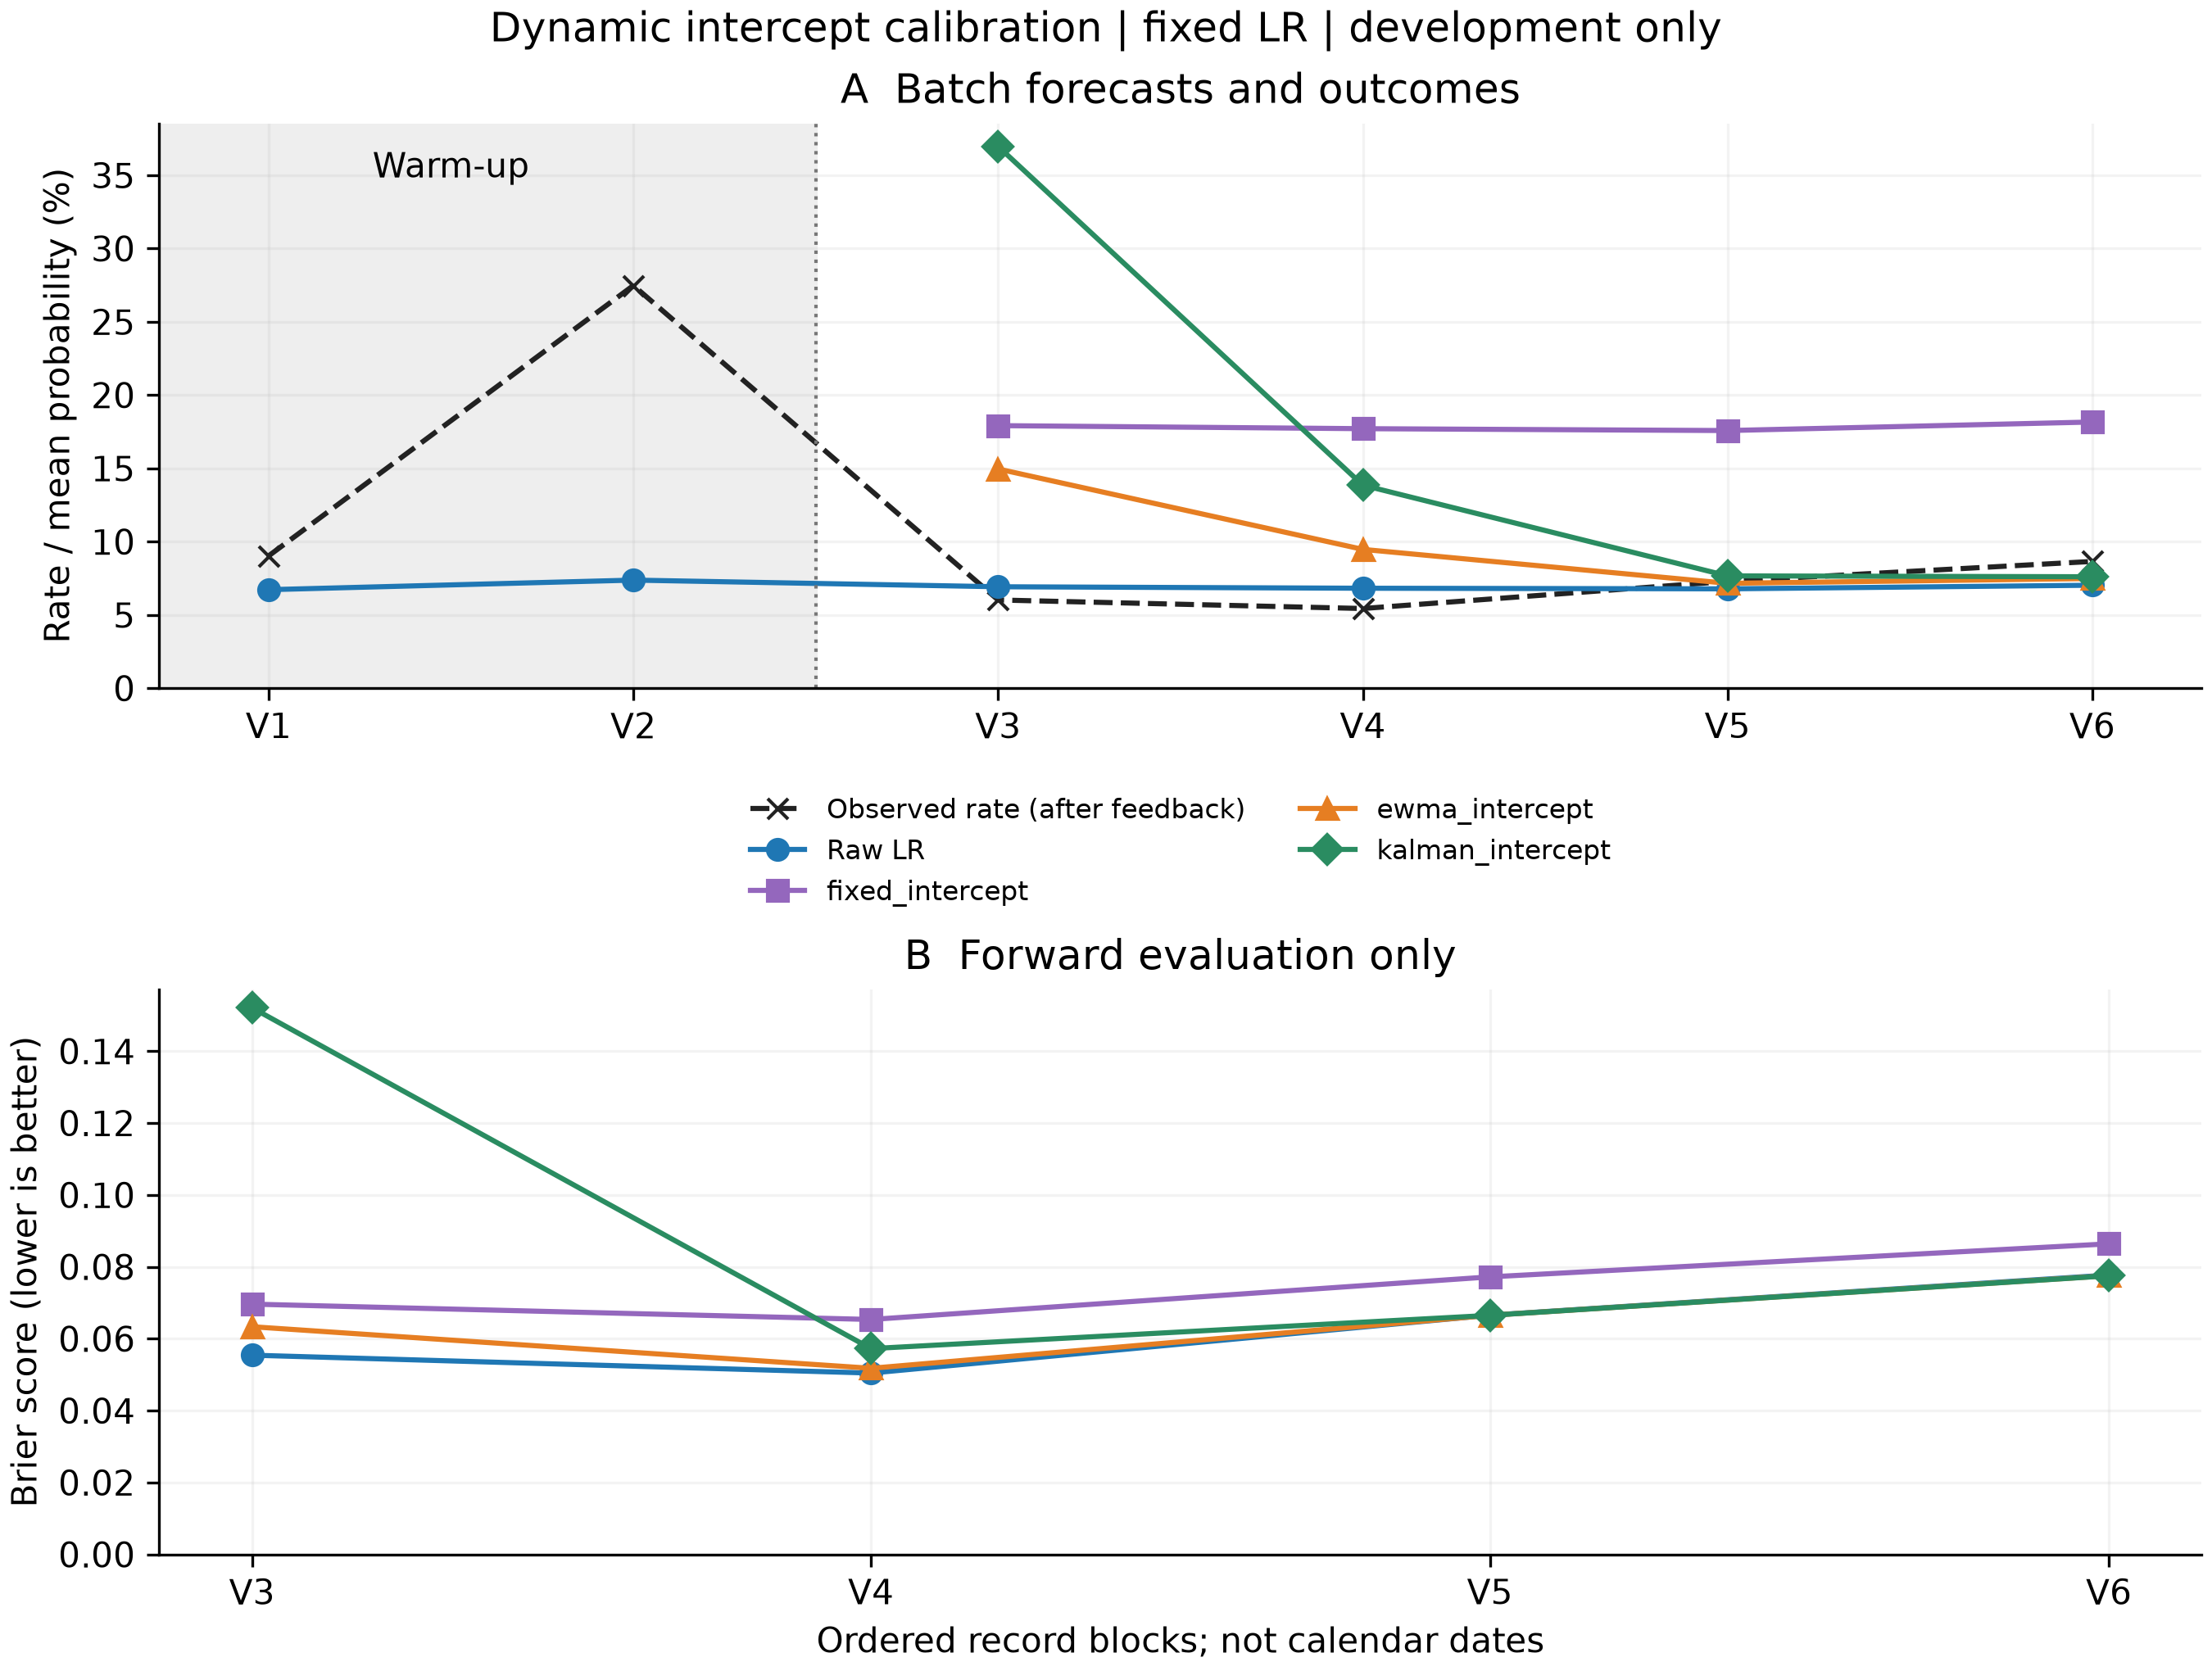

原始排序、AP、AUC、Top5/10/20名单在每块内完全不变；跨块合并排序不作区分改善证据。
只能检验概率误差是否改善，不能提高同批Top10命中。
标签在下批前全部反馈是模拟假设；缺少完整日期和成熟时间。
该记录是已见旧test后的开发探索，不能替代新未来数据的独立确认。
本cell保存实际运行结果，默认Run All不重新拟合该实验。

已完成的独立复核显示：改变当前或未来批次的标签不会影响已发出的预测。
开发阶段的完整指标见下方第9.3.1节；冻结终态后的test结果见本节主表。

#### 9.3.1 卡尔曼实验：完整指标补齐

四个方案 × V3–V6 × 四种规则，共 **64 行完整指标**；V1–V2 是预热期，不混入评价。
下表是 V3–V6 的 **逐批决策汇总**：TP/FP/FN/TN 与联系人数相加，再计算
Accuracy、Precision、Recall、F1、Lift；ROC-AUC、AP、ECE 则是先逐批计算、按批人数加权。
Brier、Log loss 和 Mean p 按人数加权，等于合并记录的对应损失和均值。
这不是四批指标的等权平均，也不是合并后重排的 Top-k；不能用这里的加权 AUC/AP 冒充 pooled AUC/AP。

**Top10% 逐批决策汇总（四组的名单相同）。**

|Model|方案|窗口|Rule|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR|raw|V3-V6|top10|4118|282|0.068480|0.627744|0.140298|0.856727|0.126214|0.184397|0.149856|0.062533|0.242281|0.012120|0.068866|412|52|360|230|3476|1.843076|
|contact_LR|ewma_intercept|V3-V6|top10|4118|282|0.068480|0.627744|0.140298|0.856727|0.126214|0.184397|0.149856|0.064792|0.254145|0.036038|0.097682|412|52|360|230|3476|1.843076|
|contact_LR|kalman_intercept|V3-V6|top10|4118|282|0.068480|0.627744|0.140298|0.856727|0.126214|0.184397|0.149856|0.088345|0.318591|0.102706|0.165255|412|52|360|230|3476|1.843076|
|contact_LR|fixed_intercept|V3-V6|top10|4118|282|0.068480|0.627744|0.140298|0.856727|0.126214|0.184397|0.149856|0.074644|0.294474|0.110523|0.178404|412|52|360|230|3476|1.843076|

**统一指标与缺失值口径。** 每行包含样本量、正例数/率、平均预测概率、ROC-AUC、AP、
Accuracy、Precision、Recall、F1、Brier、Log loss、十分箱 ECE、联系人数、TP/FP/FN/TN 和 Lift。
Top-5/10/20% 按概率降序、row_index 升序破同分，联系人数为 ceil(qN)；固定阈值为 p≥0.5。
这些是原有四种规则，不新增 F1 最优阈值搜索。概率指标使用该窗口全部记录，不随联系预算改变。

“—”表示定义不成立，不是漏算或填零：无人入选时 Precision/Lift 未定义；没有正例时
Recall/AP/Lift 未定义；单一标签时 ROC-AUC 未定义；空组的比例和损失未定义。
非空组 F1 按 zero_division=0 约定处理。分组表保留三个 poutcome 水平，
使用全窗口选出的名单与分组取交集，绝不在组内重新选 Top-k。组内 Lift 以该组正类率为基准。

原始运行文件保持不变，本次只重算保存的开发集预测，没有 fit、模型加载、新预测或原始/test 数据读取。
旧 test 已经被看过，以下仍是开发探索。原有时间加权 LR 的完整指标已在第 10 节保留。

<details>
<summary>全部 16 行逐批决策汇总；AUC/AP/ECE 为批人数加权</summary>

|Model|方案|窗口|Rule|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR|raw|V3-V6|top5|4118|282|0.068480|0.627744|0.140298|0.898009|0.168269|0.124113|0.142857|0.062533|0.242281|0.012120|0.068866|208|35|173|247|3663|2.457208|
|contact_LR|raw|V3-V6|top10|4118|282|0.068480|0.627744|0.140298|0.856727|0.126214|0.184397|0.149856|0.062533|0.242281|0.012120|0.068866|412|52|360|230|3476|1.843076|
|contact_LR|raw|V3-V6|top20|4118|282|0.068480|0.627744|0.140298|0.776591|0.112864|0.329787|0.168174|0.062533|0.242281|0.012120|0.068866|824|93|731|189|3105|1.648136|
|contact_LR|raw|V3-V6|fixed_0.5|4118|282|0.068480|0.627744|0.140298|0.931520|—|0.000000|0.000000|0.062533|0.242281|0.012120|0.068866|0|0|0|282|3836|—|
|contact_LR|ewma_intercept|V3-V6|top5|4118|282|0.068480|0.627744|0.140298|0.898009|0.168269|0.124113|0.142857|0.064792|0.254145|0.036038|0.097682|208|35|173|247|3663|2.457208|
|contact_LR|ewma_intercept|V3-V6|top10|4118|282|0.068480|0.627744|0.140298|0.856727|0.126214|0.184397|0.149856|0.064792|0.254145|0.036038|0.097682|412|52|360|230|3476|1.843076|
|contact_LR|ewma_intercept|V3-V6|top20|4118|282|0.068480|0.627744|0.140298|0.776591|0.112864|0.329787|0.168174|0.064792|0.254145|0.036038|0.097682|824|93|731|189|3105|1.648136|
|contact_LR|ewma_intercept|V3-V6|fixed_0.5|4118|282|0.068480|0.627744|0.140298|0.931520|—|0.000000|0.000000|0.064792|0.254145|0.036038|0.097682|0|0|0|282|3836|—|
|contact_LR|kalman_intercept|V3-V6|top5|4118|282|0.068480|0.627744|0.140298|0.898009|0.168269|0.124113|0.142857|0.088345|0.318591|0.102706|0.165255|208|35|173|247|3663|2.457208|
|contact_LR|kalman_intercept|V3-V6|top10|4118|282|0.068480|0.627744|0.140298|0.856727|0.126214|0.184397|0.149856|0.088345|0.318591|0.102706|0.165255|412|52|360|230|3476|1.843076|
|contact_LR|kalman_intercept|V3-V6|top20|4118|282|0.068480|0.627744|0.140298|0.776591|0.112864|0.329787|0.168174|0.088345|0.318591|0.102706|0.165255|824|93|731|189|3105|1.648136|
|contact_LR|kalman_intercept|V3-V6|fixed_0.5|4118|282|0.068480|0.627744|0.140298|0.929092|0.272727|0.021277|0.039474|0.088345|0.318591|0.102706|0.165255|22|6|16|276|3820|3.982592|
|contact_LR|fixed_intercept|V3-V6|top5|4118|282|0.068480|0.627744|0.140298|0.898009|0.168269|0.124113|0.142857|0.074644|0.294474|0.110523|0.178404|208|35|173|247|3663|2.457208|
|contact_LR|fixed_intercept|V3-V6|top10|4118|282|0.068480|0.627744|0.140298|0.856727|0.126214|0.184397|0.149856|0.074644|0.294474|0.110523|0.178404|412|52|360|230|3476|1.843076|
|contact_LR|fixed_intercept|V3-V6|top20|4118|282|0.068480|0.627744|0.140298|0.776591|0.112864|0.329787|0.168174|0.074644|0.294474|0.110523|0.178404|824|93|731|189|3105|1.648136|
|contact_LR|fixed_intercept|V3-V6|fixed_0.5|4118|282|0.068480|0.627744|0.140298|0.929577|0.357143|0.035461|0.064516|0.074644|0.294474|0.110523|0.178404|28|10|18|272|3818|5.215299|

</details>

<details>
<summary>top5：全部 16 行完整指标</summary>

|Model|方案|窗口|Rule|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR|raw|V3|top5|1030|62|0.060194|0.619943|0.136896|0.904854|0.153846|0.129032|0.140351|0.055422|0.221174|0.011421|0.069211|52|8|44|54|924|2.555831|
|contact_LR|ewma_intercept|V3|top5|1030|62|0.060194|0.619943|0.136896|0.904854|0.153846|0.129032|0.140351|0.063337|0.260212|0.089385|0.149579|52|8|44|54|924|2.555831|
|contact_LR|kalman_intercept|V3|top5|1030|62|0.060194|0.619943|0.136896|0.904854|0.153846|0.129032|0.140351|0.152077|0.491393|0.309467|0.369661|52|8|44|54|924|2.555831|
|contact_LR|fixed_intercept|V3|top5|1030|62|0.060194|0.619943|0.136896|0.904854|0.153846|0.129032|0.140351|0.069625|0.282992|0.118953|0.179148|52|8|44|54|924|2.555831|
|contact_LR|raw|V4|top5|1030|56|0.054369|0.668424|0.141210|0.908738|0.134615|0.125000|0.129630|0.050449|0.205444|0.015037|0.068202|52|7|45|49|929|2.475962|
|contact_LR|ewma_intercept|V4|top5|1030|56|0.054369|0.668424|0.141210|0.908738|0.134615|0.125000|0.129630|0.051778|0.214987|0.040339|0.094708|52|7|45|49|929|2.475962|
|contact_LR|kalman_intercept|V4|top5|1030|56|0.054369|0.668424|0.141210|0.908738|0.134615|0.125000|0.129630|0.057251|0.241571|0.084146|0.138515|52|7|45|49|929|2.475962|
|contact_LR|fixed_intercept|V4|top5|1030|56|0.054369|0.668424|0.141210|0.908738|0.134615|0.125000|0.129630|0.065354|0.271975|0.122700|0.177069|52|7|45|49|929|2.475962|
|contact_LR|raw|V5|top5|1029|75|0.072886|0.643788|0.130341|0.892128|0.153846|0.106667|0.125984|0.066554|0.253645|0.005788|0.067793|52|8|44|67|910|2.110769|
|contact_LR|ewma_intercept|V5|top5|1029|75|0.072886|0.643788|0.130341|0.892128|0.153846|0.106667|0.125984|0.066512|0.253455|0.002718|0.071555|52|8|44|67|910|2.110769|
|contact_LR|kalman_intercept|V5|top5|1029|75|0.072886|0.643788|0.130341|0.892128|0.153846|0.106667|0.125984|0.066503|0.253544|0.006575|0.076633|52|8|44|67|910|2.110769|
|contact_LR|fixed_intercept|V5|top5|1029|75|0.072886|0.643788|0.130341|0.892128|0.153846|0.106667|0.125984|0.077207|0.299099|0.104161|0.175786|52|8|44|67|910|2.110769|
|contact_LR|raw|V6|top5|1029|89|0.086492|0.578789|0.152748|0.886297|0.230769|0.134831|0.170213|0.077724|0.288917|0.016232|0.070260|52|12|40|77|900|2.668107|
|contact_LR|ewma_intercept|V6|top5|1029|89|0.086492|0.578789|0.152748|0.886297|0.230769|0.134831|0.170213|0.077555|0.287956|0.011654|0.074838|52|12|40|77|900|2.668107|
|contact_LR|kalman_intercept|V6|top5|1029|89|0.086492|0.578789|0.152748|0.886297|0.230769|0.134831|0.170213|0.077518|0.287764|0.010453|0.076039|52|12|40|77|900|2.668107|
|contact_LR|fixed_intercept|V6|top5|1029|89|0.086492|0.578789|0.152748|0.886297|0.230769|0.134831|0.170213|0.086403|0.323863|0.096258|0.181614|52|12|40|77|900|2.668107|

</details>

<details>
<summary>top10：全部 16 行完整指标</summary>

|Model|方案|窗口|Rule|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR|raw|V3|top10|1030|62|0.060194|0.619943|0.136896|0.859223|0.097087|0.161290|0.121212|0.055422|0.221174|0.011421|0.069211|103|10|93|52|875|1.612903|
|contact_LR|ewma_intercept|V3|top10|1030|62|0.060194|0.619943|0.136896|0.859223|0.097087|0.161290|0.121212|0.063337|0.260212|0.089385|0.149579|103|10|93|52|875|1.612903|
|contact_LR|kalman_intercept|V3|top10|1030|62|0.060194|0.619943|0.136896|0.859223|0.097087|0.161290|0.121212|0.152077|0.491393|0.309467|0.369661|103|10|93|52|875|1.612903|
|contact_LR|fixed_intercept|V3|top10|1030|62|0.060194|0.619943|0.136896|0.859223|0.097087|0.161290|0.121212|0.069625|0.282992|0.118953|0.179148|103|10|93|52|875|1.612903|
|contact_LR|raw|V4|top10|1030|56|0.054369|0.668424|0.141210|0.868932|0.116505|0.214286|0.150943|0.050449|0.205444|0.015037|0.068202|103|12|91|44|883|2.142857|
|contact_LR|ewma_intercept|V4|top10|1030|56|0.054369|0.668424|0.141210|0.868932|0.116505|0.214286|0.150943|0.051778|0.214987|0.040339|0.094708|103|12|91|44|883|2.142857|
|contact_LR|kalman_intercept|V4|top10|1030|56|0.054369|0.668424|0.141210|0.868932|0.116505|0.214286|0.150943|0.057251|0.241571|0.084146|0.138515|103|12|91|44|883|2.142857|
|contact_LR|fixed_intercept|V4|top10|1030|56|0.054369|0.668424|0.141210|0.868932|0.116505|0.214286|0.150943|0.065354|0.271975|0.122700|0.177069|103|12|91|44|883|2.142857|
|contact_LR|raw|V5|top10|1029|75|0.072886|0.643788|0.130341|0.858115|0.155340|0.213333|0.179775|0.066554|0.253645|0.005788|0.067793|103|16|87|59|867|2.131262|
|contact_LR|ewma_intercept|V5|top10|1029|75|0.072886|0.643788|0.130341|0.858115|0.155340|0.213333|0.179775|0.066512|0.253455|0.002718|0.071555|103|16|87|59|867|2.131262|
|contact_LR|kalman_intercept|V5|top10|1029|75|0.072886|0.643788|0.130341|0.858115|0.155340|0.213333|0.179775|0.066503|0.253544|0.006575|0.076633|103|16|87|59|867|2.131262|
|contact_LR|fixed_intercept|V5|top10|1029|75|0.072886|0.643788|0.130341|0.858115|0.155340|0.213333|0.179775|0.077207|0.299099|0.104161|0.175786|103|16|87|59|867|2.131262|
|contact_LR|raw|V6|top10|1029|89|0.086492|0.578789|0.152748|0.840622|0.135922|0.157303|0.145833|0.077724|0.288917|0.016232|0.070260|103|14|89|75|851|1.571506|
|contact_LR|ewma_intercept|V6|top10|1029|89|0.086492|0.578789|0.152748|0.840622|0.135922|0.157303|0.145833|0.077555|0.287956|0.011654|0.074838|103|14|89|75|851|1.571506|
|contact_LR|kalman_intercept|V6|top10|1029|89|0.086492|0.578789|0.152748|0.840622|0.135922|0.157303|0.145833|0.077518|0.287764|0.010453|0.076039|103|14|89|75|851|1.571506|
|contact_LR|fixed_intercept|V6|top10|1029|89|0.086492|0.578789|0.152748|0.840622|0.135922|0.157303|0.145833|0.086403|0.323863|0.096258|0.181614|103|14|89|75|851|1.571506|

</details>

<details>
<summary>top20：全部 16 行完整指标</summary>

|Model|方案|窗口|Rule|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR|raw|V3|top20|1030|62|0.060194|0.619943|0.136896|0.772816|0.082524|0.274194|0.126866|0.055422|0.221174|0.011421|0.069211|206|17|189|45|779|1.370968|
|contact_LR|ewma_intercept|V3|top20|1030|62|0.060194|0.619943|0.136896|0.772816|0.082524|0.274194|0.126866|0.063337|0.260212|0.089385|0.149579|206|17|189|45|779|1.370968|
|contact_LR|kalman_intercept|V3|top20|1030|62|0.060194|0.619943|0.136896|0.772816|0.082524|0.274194|0.126866|0.152077|0.491393|0.309467|0.369661|206|17|189|45|779|1.370968|
|contact_LR|fixed_intercept|V3|top20|1030|62|0.060194|0.619943|0.136896|0.772816|0.082524|0.274194|0.126866|0.069625|0.282992|0.118953|0.179148|206|17|189|45|779|1.370968|
|contact_LR|raw|V4|top20|1030|56|0.054369|0.668424|0.141210|0.788350|0.106796|0.392857|0.167939|0.050449|0.205444|0.015037|0.068202|206|22|184|34|790|1.964286|
|contact_LR|ewma_intercept|V4|top20|1030|56|0.054369|0.668424|0.141210|0.788350|0.106796|0.392857|0.167939|0.051778|0.214987|0.040339|0.094708|206|22|184|34|790|1.964286|
|contact_LR|kalman_intercept|V4|top20|1030|56|0.054369|0.668424|0.141210|0.788350|0.106796|0.392857|0.167939|0.057251|0.241571|0.084146|0.138515|206|22|184|34|790|1.964286|
|contact_LR|fixed_intercept|V4|top20|1030|56|0.054369|0.668424|0.141210|0.788350|0.106796|0.392857|0.167939|0.065354|0.271975|0.122700|0.177069|206|22|184|34|790|1.964286|
|contact_LR|raw|V5|top20|1029|75|0.072886|0.643788|0.130341|0.781341|0.135922|0.373333|0.199288|0.066554|0.253645|0.005788|0.067793|206|28|178|47|776|1.864854|
|contact_LR|ewma_intercept|V5|top20|1029|75|0.072886|0.643788|0.130341|0.781341|0.135922|0.373333|0.199288|0.066512|0.253455|0.002718|0.071555|206|28|178|47|776|1.864854|
|contact_LR|kalman_intercept|V5|top20|1029|75|0.072886|0.643788|0.130341|0.781341|0.135922|0.373333|0.199288|0.066503|0.253544|0.006575|0.076633|206|28|178|47|776|1.864854|
|contact_LR|fixed_intercept|V5|top20|1029|75|0.072886|0.643788|0.130341|0.781341|0.135922|0.373333|0.199288|0.077207|0.299099|0.104161|0.175786|206|28|178|47|776|1.864854|
|contact_LR|raw|V6|top20|1029|89|0.086492|0.578789|0.152748|0.763848|0.126214|0.292135|0.176271|0.077724|0.288917|0.016232|0.070260|206|26|180|63|760|1.459256|
|contact_LR|ewma_intercept|V6|top20|1029|89|0.086492|0.578789|0.152748|0.763848|0.126214|0.292135|0.176271|0.077555|0.287956|0.011654|0.074838|206|26|180|63|760|1.459256|
|contact_LR|kalman_intercept|V6|top20|1029|89|0.086492|0.578789|0.152748|0.763848|0.126214|0.292135|0.176271|0.077518|0.287764|0.010453|0.076039|206|26|180|63|760|1.459256|
|contact_LR|fixed_intercept|V6|top20|1029|89|0.086492|0.578789|0.152748|0.763848|0.126214|0.292135|0.176271|0.086403|0.323863|0.096258|0.181614|206|26|180|63|760|1.459256|

</details>

<details>
<summary>fixed_0.5：全部 16 行完整指标</summary>

|Model|方案|窗口|Rule|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR|raw|V3|fixed_0.5|1030|62|0.060194|0.619943|0.136896|0.939806|—|0.000000|0.000000|0.055422|0.221174|0.011421|0.069211|0|0|0|62|968|—|
|contact_LR|ewma_intercept|V3|fixed_0.5|1030|62|0.060194|0.619943|0.136896|0.939806|—|0.000000|0.000000|0.063337|0.260212|0.089385|0.149579|0|0|0|62|968|—|
|contact_LR|kalman_intercept|V3|fixed_0.5|1030|62|0.060194|0.619943|0.136896|0.930097|0.272727|0.096774|0.142857|0.152077|0.491393|0.309467|0.369661|22|6|16|56|952|4.530792|
|contact_LR|fixed_intercept|V3|fixed_0.5|1030|62|0.060194|0.619943|0.136896|0.937864|0.375000|0.048387|0.085714|0.069625|0.282992|0.118953|0.179148|8|3|5|59|963|6.229839|
|contact_LR|raw|V4|fixed_0.5|1030|56|0.054369|0.668424|0.141210|0.945631|—|0.000000|0.000000|0.050449|0.205444|0.015037|0.068202|0|0|0|56|974|—|
|contact_LR|ewma_intercept|V4|fixed_0.5|1030|56|0.054369|0.668424|0.141210|0.945631|—|0.000000|0.000000|0.051778|0.214987|0.040339|0.094708|0|0|0|56|974|—|
|contact_LR|kalman_intercept|V4|fixed_0.5|1030|56|0.054369|0.668424|0.141210|0.945631|—|0.000000|0.000000|0.057251|0.241571|0.084146|0.138515|0|0|0|56|974|—|
|contact_LR|fixed_intercept|V4|fixed_0.5|1030|56|0.054369|0.668424|0.141210|0.944660|0.400000|0.035714|0.065574|0.065354|0.271975|0.122700|0.177069|5|2|3|54|971|7.357143|
|contact_LR|raw|V5|fixed_0.5|1029|75|0.072886|0.643788|0.130341|0.927114|—|0.000000|0.000000|0.066554|0.253645|0.005788|0.067793|0|0|0|75|954|—|
|contact_LR|ewma_intercept|V5|fixed_0.5|1029|75|0.072886|0.643788|0.130341|0.927114|—|0.000000|0.000000|0.066512|0.253455|0.002718|0.071555|0|0|0|75|954|—|
|contact_LR|kalman_intercept|V5|fixed_0.5|1029|75|0.072886|0.643788|0.130341|0.927114|—|0.000000|0.000000|0.066503|0.253544|0.006575|0.076633|0|0|0|75|954|—|
|contact_LR|fixed_intercept|V5|fixed_0.5|1029|75|0.072886|0.643788|0.130341|0.923226|0.250000|0.026667|0.048193|0.077207|0.299099|0.104161|0.175786|8|2|6|73|948|3.430000|
|contact_LR|raw|V6|fixed_0.5|1029|89|0.086492|0.578789|0.152748|0.913508|—|0.000000|0.000000|0.077724|0.288917|0.016232|0.070260|0|0|0|89|940|—|
|contact_LR|ewma_intercept|V6|fixed_0.5|1029|89|0.086492|0.578789|0.152748|0.913508|—|0.000000|0.000000|0.077555|0.287956|0.011654|0.074838|0|0|0|89|940|—|
|contact_LR|kalman_intercept|V6|fixed_0.5|1029|89|0.086492|0.578789|0.152748|0.913508|—|0.000000|0.000000|0.077518|0.287764|0.010453|0.076039|0|0|0|89|940|—|
|contact_LR|fixed_intercept|V6|fixed_0.5|1029|89|0.086492|0.578789|0.152748|0.912536|0.428571|0.033708|0.062500|0.086403|0.323863|0.096258|0.181614|7|3|4|86|936|4.955056|

</details>

<details>
<summary>top5：poutcome 分组完整指标，共 48 行</summary>

|Model|方案|窗口|Rule|poutcome|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR|raw|V3|top5|nonexistent|663|41|0.061840|0.589954|0.077943|0.900452|0.068966|0.048780|0.057143|0.057837|0.230273|0.006672|0.068512|29|2|27|39|595|1.115223|
|contact_LR|raw|V3|top5|failure|346|15|0.043353|0.556596|0.049701|0.947977|0.000000|0.000000|0.000000|0.041799|0.180911|0.017661|0.061013|3|0|3|15|328|0.000000|
|contact_LR|raw|V3|top5|success|21|6|0.285714|0.622222|0.594139|0.333333|0.300000|1.000000|0.461538|0.203647|0.597266|0.067013|0.226337|20|6|14|0|1|1.050000|
|contact_LR|ewma_intercept|V3|top5|nonexistent|663|41|0.061840|0.589954|0.077943|0.900452|0.068966|0.048780|0.057143|0.065491|0.267383|0.087514|0.149355|29|2|27|39|595|1.115223|
|contact_LR|ewma_intercept|V3|top5|failure|346|15|0.043353|0.556596|0.049701|0.947977|0.000000|0.000000|0.000000|0.049988|0.224594|0.090964|0.134317|3|0|3|15|328|0.000000|
|contact_LR|ewma_intercept|V3|top5|success|21|6|0.285714|0.622222|0.594139|0.333333|0.300000|1.000000|0.461538|0.215289|0.620666|0.122412|0.408126|20|6|14|0|1|1.050000|
|contact_LR|kalman_intercept|V3|top5|nonexistent|663|41|0.061840|0.589954|0.077943|0.900452|0.068966|0.048780|0.057143|0.155057|0.497955|0.310751|0.372591|29|2|27|39|595|1.115223|
|contact_LR|kalman_intercept|V3|top5|failure|346|15|0.043353|0.556596|0.049701|0.947977|0.000000|0.000000|0.000000|0.133248|0.450953|0.300958|0.344310|3|0|3|15|328|0.000000|
|contact_LR|kalman_intercept|V3|top5|success|21|6|0.285714|0.622222|0.594139|0.333333|0.300000|1.000000|0.461538|0.368217|0.950519|0.409140|0.694854|20|6|14|0|1|1.050000|
|contact_LR|fixed_intercept|V3|top5|nonexistent|663|41|0.061840|0.589954|0.077943|0.900452|0.068966|0.048780|0.057143|0.071690|0.289789|0.117435|0.179275|29|2|27|39|595|1.115223|
|contact_LR|fixed_intercept|V3|top5|failure|346|15|0.043353|0.556596|0.049701|0.947977|0.000000|0.000000|0.000000|0.055866|0.247493|0.118459|0.161811|3|0|3|15|328|0.000000|
|contact_LR|fixed_intercept|V3|top5|success|21|6|0.285714|0.622222|0.594139|0.333333|0.300000|1.000000|0.461538|0.231147|0.653275|0.175043|0.460757|20|6|14|0|1|1.050000|
|contact_LR|raw|V4|top5|nonexistent|673|42|0.062407|0.615821|0.095773|0.898960|0.093750|0.071429|0.081081|0.058144|0.230388|0.005373|0.067780|32|3|29|39|602|1.502232|
|contact_LR|raw|V4|top5|failure|340|10|0.029412|0.698788|0.075531|0.961765|0.000000|0.000000|0.000000|0.029405|0.141070|0.032144|0.061555|3|0|3|10|327|0.000000|
|contact_LR|raw|V4|top5|success|17|4|0.235294|0.750000|0.674242|0.235294|0.235294|1.000000|0.380952|0.166651|0.505457|0.081785|0.217852|17|4|13|0|0|1.000000|
|contact_LR|ewma_intercept|V4|top5|nonexistent|673|42|0.062407|0.615821|0.095773|0.898960|0.093750|0.071429|0.081081|0.059077|0.236888|0.031964|0.094371|32|3|29|39|602|1.502232|
|contact_LR|ewma_intercept|V4|top5|failure|340|10|0.029412|0.698788|0.075531|0.961765|0.000000|0.000000|0.000000|0.031580|0.156847|0.056494|0.085905|3|0|3|10|327|0.000000|
|contact_LR|ewma_intercept|V4|top5|success|17|4|0.235294|0.750000|0.674242|0.235294|0.235294|1.000000|0.380952|0.166805|0.510777|0.058828|0.284110|17|4|13|0|0|1.000000|
|contact_LR|kalman_intercept|V4|top5|nonexistent|673|42|0.062407|0.615821|0.095773|0.898960|0.093750|0.071429|0.081081|0.063834|0.259884|0.076092|0.138499|32|3|29|39|602|1.502232|
|contact_LR|kalman_intercept|V4|top5|failure|340|10|0.029412|0.698788|0.075531|0.961765|0.000000|0.000000|0.000000|0.037925|0.189802|0.097172|0.126584|3|0|3|10|327|0.000000|
|contact_LR|kalman_intercept|V4|top5|success|17|4|0.235294|0.750000|0.674242|0.235294|0.235294|1.000000|0.380952|0.183158|0.551951|0.142475|0.377769|17|4|13|0|0|1.000000|
|contact_LR|fixed_intercept|V4|top5|nonexistent|673|42|0.062407|0.615821|0.095773|0.898960|0.093750|0.071429|0.081081|0.071342|0.287961|0.115049|0.177456|32|3|29|39|602|1.502232|
|contact_LR|fixed_intercept|V4|top5|failure|340|10|0.029412|0.698788|0.075531|0.961765|0.000000|0.000000|0.000000|0.046402|0.223715|0.133375|0.162787|3|0|3|10|327|0.000000|
|contact_LR|fixed_intercept|V4|top5|success|17|4|0.235294|0.750000|0.674242|0.235294|0.235294|1.000000|0.380952|0.207353|0.604307|0.212080|0.447374|17|4|13|0|0|1.000000|
|contact_LR|raw|V5|top5|nonexistent|670|55|0.082090|0.631648|0.118247|0.877612|0.064516|0.036364|0.046512|0.074831|0.279278|0.015324|0.067263|31|2|29|53|586|0.785924|
|contact_LR|raw|V5|top5|failure|341|15|0.043988|0.532209|0.079031|0.953079|0.333333|0.066667|0.111111|0.042497|0.182766|0.016920|0.060909|3|1|2|14|324|7.577778|
|contact_LR|raw|V5|top5|success|18|5|0.277778|0.461538|0.322222|0.277778|0.277778|1.000000|0.434783|0.214216|0.642268|0.065743|0.217947|18|5|13|0|0|1.000000|
|contact_LR|ewma_intercept|V5|top5|nonexistent|670|55|0.082090|0.631648|0.118247|0.877612|0.064516|0.036364|0.046512|0.074706|0.278517|0.012358|0.071029|31|2|29|53|586|0.785924|
|contact_LR|ewma_intercept|V5|top5|failure|341|15|0.043988|0.532209|0.079031|0.953079|0.333333|0.066667|0.111111|0.042645|0.183860|0.025016|0.064335|3|1|2|14|324|7.577778|
|contact_LR|ewma_intercept|V5|top5|success|18|5|0.277778|0.461538|0.322222|0.277778|0.277778|1.000000|0.434783|0.213653|0.639044|0.093945|0.227895|18|5|13|0|0|1.000000|
|contact_LR|kalman_intercept|V5|top5|nonexistent|670|55|0.082090|0.631648|0.118247|0.877612|0.064516|0.036364|0.046512|0.074583|0.277877|0.008298|0.076118|31|2|29|53|586|0.785924|
|contact_LR|kalman_intercept|V5|top5|failure|341|15|0.043988|0.532209|0.079031|0.953079|0.333333|0.066667|0.111111|0.042883|0.185556|0.029565|0.068967|3|1|2|14|324|7.577778|
|contact_LR|kalman_intercept|V5|top5|success|18|5|0.277778|0.461538|0.322222|0.277778|0.277778|1.000000|0.434783|0.213210|0.635795|0.124631|0.241033|18|5|13|0|0|1.000000|
|contact_LR|fixed_intercept|V5|top5|nonexistent|670|55|0.082090|0.631648|0.118247|0.877612|0.064516|0.036364|0.046512|0.083066|0.314398|0.094031|0.176121|31|2|29|53|586|0.785924|
|contact_LR|fixed_intercept|V5|top5|failure|341|15|0.043988|0.532209|0.079031|0.953079|0.333333|0.066667|0.111111|0.056620|0.248190|0.116884|0.160872|3|1|2|14|324|7.577778|
|contact_LR|fixed_intercept|V5|top5|success|18|5|0.277778|0.461538|0.322222|0.277778|0.277778|1.000000|0.434783|0.249137|0.694082|0.260781|0.445846|18|5|13|0|0|1.000000|
|contact_LR|raw|V6|top5|nonexistent|701|61|0.087019|0.546568|0.106523|0.883024|0.161290|0.081967|0.108696|0.079590|0.296974|0.017957|0.069061|31|5|26|56|614|1.853517|
|contact_LR|raw|V6|top5|failure|312|22|0.070513|0.560266|0.128820|0.916667|0.166667|0.045455|0.071429|0.064276|0.248684|0.006583|0.064990|6|1|5|21|285|2.363636|
|contact_LR|raw|V6|top5|success|16|6|0.375000|0.450000|0.378677|0.437500|0.400000|1.000000|0.571429|0.258177|0.720442|0.158153|0.225532|15|6|9|0|1|1.066667|
|contact_LR|ewma_intercept|V6|top5|nonexistent|701|61|0.087019|0.546568|0.106523|0.883024|0.161290|0.081967|0.108696|0.079449|0.295894|0.013417|0.073602|31|5|26|56|614|1.853517|
|contact_LR|ewma_intercept|V6|top5|failure|312|22|0.070513|0.560266|0.128820|0.916667|0.166667|0.045455|0.071429|0.064207|0.248450|0.003685|0.069269|6|1|5|21|285|2.363636|
|contact_LR|ewma_intercept|V6|top5|success|16|6|0.375000|0.450000|0.378677|0.437500|0.400000|1.000000|0.571429|0.254833|0.710573|0.185080|0.237558|15|6|9|0|1|1.066667|
|contact_LR|kalman_intercept|V6|top5|nonexistent|701|61|0.087019|0.546568|0.106523|0.883024|0.161290|0.081967|0.108696|0.079420|0.295670|0.012224|0.074794|31|5|26|56|614|1.853517|
|contact_LR|kalman_intercept|V6|top5|failure|312|22|0.070513|0.560266|0.128820|0.916667|0.166667|0.045455|0.071429|0.064196|0.248438|0.004280|0.070393|6|1|5|21|285|2.363636|
|contact_LR|kalman_intercept|V6|top5|success|16|6|0.375000|0.450000|0.378677|0.437500|0.400000|1.000000|0.571429|0.254015|0.708206|0.220192|0.240670|15|6|9|0|1|1.066667|
|contact_LR|fixed_intercept|V6|top5|nonexistent|701|61|0.087019|0.546568|0.106523|0.883024|0.161290|0.081967|0.108696|0.088333|0.329861|0.095618|0.180316|31|5|26|56|614|1.853517|
|contact_LR|fixed_intercept|V6|top5|failure|312|22|0.070513|0.560266|0.128820|0.916667|0.166667|0.045455|0.071429|0.073995|0.292267|0.102681|0.170345|6|1|5|21|285|2.363636|
|contact_LR|fixed_intercept|V6|top5|success|16|6|0.375000|0.450000|0.378677|0.437500|0.400000|1.000000|0.571429|0.243813|0.677219|0.135567|0.458251|15|6|9|0|1|1.066667|

</details>

<details>
<summary>top10：poutcome 分组完整指标，共 48 行</summary>

|Model|方案|窗口|Rule|poutcome|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR|raw|V3|top10|nonexistent|663|41|0.061840|0.589954|0.077943|0.843137|0.056338|0.097561|0.071429|0.057837|0.230273|0.006672|0.068512|71|4|67|37|555|0.911027|
|contact_LR|raw|V3|top10|failure|346|15|0.043353|0.556596|0.049701|0.921965|0.000000|0.000000|0.000000|0.041799|0.180911|0.017661|0.061013|12|0|12|15|319|0.000000|
|contact_LR|raw|V3|top10|success|21|6|0.285714|0.622222|0.594139|0.333333|0.300000|1.000000|0.461538|0.203647|0.597266|0.067013|0.226337|20|6|14|0|1|1.050000|
|contact_LR|ewma_intercept|V3|top10|nonexistent|663|41|0.061840|0.589954|0.077943|0.843137|0.056338|0.097561|0.071429|0.065491|0.267383|0.087514|0.149355|71|4|67|37|555|0.911027|
|contact_LR|ewma_intercept|V3|top10|failure|346|15|0.043353|0.556596|0.049701|0.921965|0.000000|0.000000|0.000000|0.049988|0.224594|0.090964|0.134317|12|0|12|15|319|0.000000|
|contact_LR|ewma_intercept|V3|top10|success|21|6|0.285714|0.622222|0.594139|0.333333|0.300000|1.000000|0.461538|0.215289|0.620666|0.122412|0.408126|20|6|14|0|1|1.050000|
|contact_LR|kalman_intercept|V3|top10|nonexistent|663|41|0.061840|0.589954|0.077943|0.843137|0.056338|0.097561|0.071429|0.155057|0.497955|0.310751|0.372591|71|4|67|37|555|0.911027|
|contact_LR|kalman_intercept|V3|top10|failure|346|15|0.043353|0.556596|0.049701|0.921965|0.000000|0.000000|0.000000|0.133248|0.450953|0.300958|0.344310|12|0|12|15|319|0.000000|
|contact_LR|kalman_intercept|V3|top10|success|21|6|0.285714|0.622222|0.594139|0.333333|0.300000|1.000000|0.461538|0.368217|0.950519|0.409140|0.694854|20|6|14|0|1|1.050000|
|contact_LR|fixed_intercept|V3|top10|nonexistent|663|41|0.061840|0.589954|0.077943|0.843137|0.056338|0.097561|0.071429|0.071690|0.289789|0.117435|0.179275|71|4|67|37|555|0.911027|
|contact_LR|fixed_intercept|V3|top10|failure|346|15|0.043353|0.556596|0.049701|0.921965|0.000000|0.000000|0.000000|0.055866|0.247493|0.118459|0.161811|12|0|12|15|319|0.000000|
|contact_LR|fixed_intercept|V3|top10|success|21|6|0.285714|0.622222|0.594139|0.333333|0.300000|1.000000|0.461538|0.231147|0.653275|0.175043|0.460757|20|6|14|0|1|1.050000|
|contact_LR|raw|V4|top10|nonexistent|673|42|0.062407|0.615821|0.095773|0.843982|0.101266|0.190476|0.132231|0.058144|0.230388|0.005373|0.067780|79|8|71|34|560|1.622664|
|contact_LR|raw|V4|top10|failure|340|10|0.029412|0.698788|0.075531|0.950000|0.000000|0.000000|0.000000|0.029405|0.141070|0.032144|0.061555|7|0|7|10|323|0.000000|
|contact_LR|raw|V4|top10|success|17|4|0.235294|0.750000|0.674242|0.235294|0.235294|1.000000|0.380952|0.166651|0.505457|0.081785|0.217852|17|4|13|0|0|1.000000|
|contact_LR|ewma_intercept|V4|top10|nonexistent|673|42|0.062407|0.615821|0.095773|0.843982|0.101266|0.190476|0.132231|0.059077|0.236888|0.031964|0.094371|79|8|71|34|560|1.622664|
|contact_LR|ewma_intercept|V4|top10|failure|340|10|0.029412|0.698788|0.075531|0.950000|0.000000|0.000000|0.000000|0.031580|0.156847|0.056494|0.085905|7|0|7|10|323|0.000000|
|contact_LR|ewma_intercept|V4|top10|success|17|4|0.235294|0.750000|0.674242|0.235294|0.235294|1.000000|0.380952|0.166805|0.510777|0.058828|0.284110|17|4|13|0|0|1.000000|
|contact_LR|kalman_intercept|V4|top10|nonexistent|673|42|0.062407|0.615821|0.095773|0.843982|0.101266|0.190476|0.132231|0.063834|0.259884|0.076092|0.138499|79|8|71|34|560|1.622664|
|contact_LR|kalman_intercept|V4|top10|failure|340|10|0.029412|0.698788|0.075531|0.950000|0.000000|0.000000|0.000000|0.037925|0.189802|0.097172|0.126584|7|0|7|10|323|0.000000|
|contact_LR|kalman_intercept|V4|top10|success|17|4|0.235294|0.750000|0.674242|0.235294|0.235294|1.000000|0.380952|0.183158|0.551951|0.142475|0.377769|17|4|13|0|0|1.000000|
|contact_LR|fixed_intercept|V4|top10|nonexistent|673|42|0.062407|0.615821|0.095773|0.843982|0.101266|0.190476|0.132231|0.071342|0.287961|0.115049|0.177456|79|8|71|34|560|1.622664|
|contact_LR|fixed_intercept|V4|top10|failure|340|10|0.029412|0.698788|0.075531|0.950000|0.000000|0.000000|0.000000|0.046402|0.223715|0.133375|0.162787|7|0|7|10|323|0.000000|
|contact_LR|fixed_intercept|V4|top10|success|17|4|0.235294|0.750000|0.674242|0.235294|0.235294|1.000000|0.380952|0.207353|0.604307|0.212080|0.447374|17|4|13|0|0|1.000000|
|contact_LR|raw|V5|top10|nonexistent|670|55|0.082090|0.631648|0.118247|0.829851|0.126582|0.181818|0.149254|0.074831|0.279278|0.015324|0.067263|79|10|69|45|546|1.542002|
|contact_LR|raw|V5|top10|failure|341|15|0.043988|0.532209|0.079031|0.944282|0.166667|0.066667|0.095238|0.042497|0.182766|0.016920|0.060909|6|1|5|14|321|3.788889|
|contact_LR|raw|V5|top10|success|18|5|0.277778|0.461538|0.322222|0.277778|0.277778|1.000000|0.434783|0.214216|0.642268|0.065743|0.217947|18|5|13|0|0|1.000000|
|contact_LR|ewma_intercept|V5|top10|nonexistent|670|55|0.082090|0.631648|0.118247|0.829851|0.126582|0.181818|0.149254|0.074706|0.278517|0.012358|0.071029|79|10|69|45|546|1.542002|
|contact_LR|ewma_intercept|V5|top10|failure|341|15|0.043988|0.532209|0.079031|0.944282|0.166667|0.066667|0.095238|0.042645|0.183860|0.025016|0.064335|6|1|5|14|321|3.788889|
|contact_LR|ewma_intercept|V5|top10|success|18|5|0.277778|0.461538|0.322222|0.277778|0.277778|1.000000|0.434783|0.213653|0.639044|0.093945|0.227895|18|5|13|0|0|1.000000|
|contact_LR|kalman_intercept|V5|top10|nonexistent|670|55|0.082090|0.631648|0.118247|0.829851|0.126582|0.181818|0.149254|0.074583|0.277877|0.008298|0.076118|79|10|69|45|546|1.542002|
|contact_LR|kalman_intercept|V5|top10|failure|341|15|0.043988|0.532209|0.079031|0.944282|0.166667|0.066667|0.095238|0.042883|0.185556|0.029565|0.068967|6|1|5|14|321|3.788889|
|contact_LR|kalman_intercept|V5|top10|success|18|5|0.277778|0.461538|0.322222|0.277778|0.277778|1.000000|0.434783|0.213210|0.635795|0.124631|0.241033|18|5|13|0|0|1.000000|
|contact_LR|fixed_intercept|V5|top10|nonexistent|670|55|0.082090|0.631648|0.118247|0.829851|0.126582|0.181818|0.149254|0.083066|0.314398|0.094031|0.176121|79|10|69|45|546|1.542002|
|contact_LR|fixed_intercept|V5|top10|failure|341|15|0.043988|0.532209|0.079031|0.944282|0.166667|0.066667|0.095238|0.056620|0.248190|0.116884|0.160872|6|1|5|14|321|3.788889|
|contact_LR|fixed_intercept|V5|top10|success|18|5|0.277778|0.461538|0.322222|0.277778|0.277778|1.000000|0.434783|0.249137|0.694082|0.260781|0.445846|18|5|13|0|0|1.000000|
|contact_LR|raw|V6|top10|nonexistent|701|61|0.087019|0.546568|0.106523|0.821683|0.078947|0.098361|0.087591|0.079590|0.296974|0.017957|0.069061|76|6|70|55|570|0.907248|
|contact_LR|raw|V6|top10|failure|312|22|0.070513|0.560266|0.128820|0.903846|0.166667|0.090909|0.117647|0.064276|0.248684|0.006583|0.064990|12|2|10|20|280|2.363636|
|contact_LR|raw|V6|top10|success|16|6|0.375000|0.450000|0.378677|0.437500|0.400000|1.000000|0.571429|0.258177|0.720442|0.158153|0.225532|15|6|9|0|1|1.066667|
|contact_LR|ewma_intercept|V6|top10|nonexistent|701|61|0.087019|0.546568|0.106523|0.821683|0.078947|0.098361|0.087591|0.079449|0.295894|0.013417|0.073602|76|6|70|55|570|0.907248|
|contact_LR|ewma_intercept|V6|top10|failure|312|22|0.070513|0.560266|0.128820|0.903846|0.166667|0.090909|0.117647|0.064207|0.248450|0.003685|0.069269|12|2|10|20|280|2.363636|
|contact_LR|ewma_intercept|V6|top10|success|16|6|0.375000|0.450000|0.378677|0.437500|0.400000|1.000000|0.571429|0.254833|0.710573|0.185080|0.237558|15|6|9|0|1|1.066667|
|contact_LR|kalman_intercept|V6|top10|nonexistent|701|61|0.087019|0.546568|0.106523|0.821683|0.078947|0.098361|0.087591|0.079420|0.295670|0.012224|0.074794|76|6|70|55|570|0.907248|
|contact_LR|kalman_intercept|V6|top10|failure|312|22|0.070513|0.560266|0.128820|0.903846|0.166667|0.090909|0.117647|0.064196|0.248438|0.004280|0.070393|12|2|10|20|280|2.363636|
|contact_LR|kalman_intercept|V6|top10|success|16|6|0.375000|0.450000|0.378677|0.437500|0.400000|1.000000|0.571429|0.254015|0.708206|0.220192|0.240670|15|6|9|0|1|1.066667|
|contact_LR|fixed_intercept|V6|top10|nonexistent|701|61|0.087019|0.546568|0.106523|0.821683|0.078947|0.098361|0.087591|0.088333|0.329861|0.095618|0.180316|76|6|70|55|570|0.907248|
|contact_LR|fixed_intercept|V6|top10|failure|312|22|0.070513|0.560266|0.128820|0.903846|0.166667|0.090909|0.117647|0.073995|0.292267|0.102681|0.170345|12|2|10|20|280|2.363636|
|contact_LR|fixed_intercept|V6|top10|success|16|6|0.375000|0.450000|0.378677|0.437500|0.400000|1.000000|0.571429|0.243813|0.677219|0.135567|0.458251|15|6|9|0|1|1.066667|

</details>

<details>
<summary>top20：poutcome 分组完整指标，共 48 行</summary>

|Model|方案|窗口|Rule|poutcome|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR|raw|V3|top20|nonexistent|663|41|0.061840|0.589954|0.077943|0.737557|0.070968|0.268293|0.112245|0.057837|0.230273|0.006672|0.068512|155|11|144|30|478|1.147600|
|contact_LR|raw|V3|top20|failure|346|15|0.043353|0.556596|0.049701|0.869942|0.000000|0.000000|0.000000|0.041799|0.180911|0.017661|0.061013|30|0|30|15|301|0.000000|
|contact_LR|raw|V3|top20|success|21|6|0.285714|0.622222|0.594139|0.285714|0.285714|1.000000|0.444444|0.203647|0.597266|0.067013|0.226337|21|6|15|0|0|1.000000|
|contact_LR|ewma_intercept|V3|top20|nonexistent|663|41|0.061840|0.589954|0.077943|0.737557|0.070968|0.268293|0.112245|0.065491|0.267383|0.087514|0.149355|155|11|144|30|478|1.147600|
|contact_LR|ewma_intercept|V3|top20|failure|346|15|0.043353|0.556596|0.049701|0.869942|0.000000|0.000000|0.000000|0.049988|0.224594|0.090964|0.134317|30|0|30|15|301|0.000000|
|contact_LR|ewma_intercept|V3|top20|success|21|6|0.285714|0.622222|0.594139|0.285714|0.285714|1.000000|0.444444|0.215289|0.620666|0.122412|0.408126|21|6|15|0|0|1.000000|
|contact_LR|kalman_intercept|V3|top20|nonexistent|663|41|0.061840|0.589954|0.077943|0.737557|0.070968|0.268293|0.112245|0.155057|0.497955|0.310751|0.372591|155|11|144|30|478|1.147600|
|contact_LR|kalman_intercept|V3|top20|failure|346|15|0.043353|0.556596|0.049701|0.869942|0.000000|0.000000|0.000000|0.133248|0.450953|0.300958|0.344310|30|0|30|15|301|0.000000|
|contact_LR|kalman_intercept|V3|top20|success|21|6|0.285714|0.622222|0.594139|0.285714|0.285714|1.000000|0.444444|0.368217|0.950519|0.409140|0.694854|21|6|15|0|0|1.000000|
|contact_LR|fixed_intercept|V3|top20|nonexistent|663|41|0.061840|0.589954|0.077943|0.737557|0.070968|0.268293|0.112245|0.071690|0.289789|0.117435|0.179275|155|11|144|30|478|1.147600|
|contact_LR|fixed_intercept|V3|top20|failure|346|15|0.043353|0.556596|0.049701|0.869942|0.000000|0.000000|0.000000|0.055866|0.247493|0.118459|0.161811|30|0|30|15|301|0.000000|
|contact_LR|fixed_intercept|V3|top20|success|21|6|0.285714|0.622222|0.594139|0.285714|0.285714|1.000000|0.444444|0.231147|0.653275|0.175043|0.460757|21|6|15|0|0|1.000000|
|contact_LR|raw|V4|top20|nonexistent|673|42|0.062407|0.615821|0.095773|0.745914|0.094340|0.357143|0.149254|0.058144|0.230388|0.005373|0.067780|159|15|144|27|487|1.511680|
|contact_LR|raw|V4|top20|failure|340|10|0.029412|0.698788|0.075531|0.900000|0.100000|0.300000|0.150000|0.029405|0.141070|0.032144|0.061555|30|3|27|7|303|3.400000|
|contact_LR|raw|V4|top20|success|17|4|0.235294|0.750000|0.674242|0.235294|0.235294|1.000000|0.380952|0.166651|0.505457|0.081785|0.217852|17|4|13|0|0|1.000000|
|contact_LR|ewma_intercept|V4|top20|nonexistent|673|42|0.062407|0.615821|0.095773|0.745914|0.094340|0.357143|0.149254|0.059077|0.236888|0.031964|0.094371|159|15|144|27|487|1.511680|
|contact_LR|ewma_intercept|V4|top20|failure|340|10|0.029412|0.698788|0.075531|0.900000|0.100000|0.300000|0.150000|0.031580|0.156847|0.056494|0.085905|30|3|27|7|303|3.400000|
|contact_LR|ewma_intercept|V4|top20|success|17|4|0.235294|0.750000|0.674242|0.235294|0.235294|1.000000|0.380952|0.166805|0.510777|0.058828|0.284110|17|4|13|0|0|1.000000|
|contact_LR|kalman_intercept|V4|top20|nonexistent|673|42|0.062407|0.615821|0.095773|0.745914|0.094340|0.357143|0.149254|0.063834|0.259884|0.076092|0.138499|159|15|144|27|487|1.511680|
|contact_LR|kalman_intercept|V4|top20|failure|340|10|0.029412|0.698788|0.075531|0.900000|0.100000|0.300000|0.150000|0.037925|0.189802|0.097172|0.126584|30|3|27|7|303|3.400000|
|contact_LR|kalman_intercept|V4|top20|success|17|4|0.235294|0.750000|0.674242|0.235294|0.235294|1.000000|0.380952|0.183158|0.551951|0.142475|0.377769|17|4|13|0|0|1.000000|
|contact_LR|fixed_intercept|V4|top20|nonexistent|673|42|0.062407|0.615821|0.095773|0.745914|0.094340|0.357143|0.149254|0.071342|0.287961|0.115049|0.177456|159|15|144|27|487|1.511680|
|contact_LR|fixed_intercept|V4|top20|failure|340|10|0.029412|0.698788|0.075531|0.900000|0.100000|0.300000|0.150000|0.046402|0.223715|0.133375|0.162787|30|3|27|7|303|3.400000|
|contact_LR|fixed_intercept|V4|top20|success|17|4|0.235294|0.750000|0.674242|0.235294|0.235294|1.000000|0.380952|0.207353|0.604307|0.212080|0.447374|17|4|13|0|0|1.000000|
|contact_LR|raw|V5|top20|nonexistent|670|55|0.082090|0.631648|0.118247|0.746269|0.138365|0.400000|0.205607|0.074831|0.279278|0.015324|0.067263|159|22|137|33|478|1.685535|
|contact_LR|raw|V5|top20|failure|341|15|0.043988|0.532209|0.079031|0.876833|0.034483|0.066667|0.045455|0.042497|0.182766|0.016920|0.060909|29|1|28|14|298|0.783908|
|contact_LR|raw|V5|top20|success|18|5|0.277778|0.461538|0.322222|0.277778|0.277778|1.000000|0.434783|0.214216|0.642268|0.065743|0.217947|18|5|13|0|0|1.000000|
|contact_LR|ewma_intercept|V5|top20|nonexistent|670|55|0.082090|0.631648|0.118247|0.746269|0.138365|0.400000|0.205607|0.074706|0.278517|0.012358|0.071029|159|22|137|33|478|1.685535|
|contact_LR|ewma_intercept|V5|top20|failure|341|15|0.043988|0.532209|0.079031|0.876833|0.034483|0.066667|0.045455|0.042645|0.183860|0.025016|0.064335|29|1|28|14|298|0.783908|
|contact_LR|ewma_intercept|V5|top20|success|18|5|0.277778|0.461538|0.322222|0.277778|0.277778|1.000000|0.434783|0.213653|0.639044|0.093945|0.227895|18|5|13|0|0|1.000000|
|contact_LR|kalman_intercept|V5|top20|nonexistent|670|55|0.082090|0.631648|0.118247|0.746269|0.138365|0.400000|0.205607|0.074583|0.277877|0.008298|0.076118|159|22|137|33|478|1.685535|
|contact_LR|kalman_intercept|V5|top20|failure|341|15|0.043988|0.532209|0.079031|0.876833|0.034483|0.066667|0.045455|0.042883|0.185556|0.029565|0.068967|29|1|28|14|298|0.783908|
|contact_LR|kalman_intercept|V5|top20|success|18|5|0.277778|0.461538|0.322222|0.277778|0.277778|1.000000|0.434783|0.213210|0.635795|0.124631|0.241033|18|5|13|0|0|1.000000|
|contact_LR|fixed_intercept|V5|top20|nonexistent|670|55|0.082090|0.631648|0.118247|0.746269|0.138365|0.400000|0.205607|0.083066|0.314398|0.094031|0.176121|159|22|137|33|478|1.685535|
|contact_LR|fixed_intercept|V5|top20|failure|341|15|0.043988|0.532209|0.079031|0.876833|0.034483|0.066667|0.045455|0.056620|0.248190|0.116884|0.160872|29|1|28|14|298|0.783908|
|contact_LR|fixed_intercept|V5|top20|success|18|5|0.277778|0.461538|0.322222|0.277778|0.277778|1.000000|0.434783|0.249137|0.694082|0.260781|0.445846|18|5|13|0|0|1.000000|
|contact_LR|raw|V6|top20|nonexistent|701|61|0.087019|0.546568|0.106523|0.743224|0.111111|0.278689|0.158879|0.079590|0.296974|0.017957|0.069061|153|17|136|44|504|1.276867|
|contact_LR|raw|V6|top20|failure|312|22|0.070513|0.560266|0.128820|0.826923|0.078947|0.136364|0.100000|0.064276|0.248684|0.006583|0.064990|38|3|35|19|255|1.119617|
|contact_LR|raw|V6|top20|success|16|6|0.375000|0.450000|0.378677|0.437500|0.400000|1.000000|0.571429|0.258177|0.720442|0.158153|0.225532|15|6|9|0|1|1.066667|
|contact_LR|ewma_intercept|V6|top20|nonexistent|701|61|0.087019|0.546568|0.106523|0.743224|0.111111|0.278689|0.158879|0.079449|0.295894|0.013417|0.073602|153|17|136|44|504|1.276867|
|contact_LR|ewma_intercept|V6|top20|failure|312|22|0.070513|0.560266|0.128820|0.826923|0.078947|0.136364|0.100000|0.064207|0.248450|0.003685|0.069269|38|3|35|19|255|1.119617|
|contact_LR|ewma_intercept|V6|top20|success|16|6|0.375000|0.450000|0.378677|0.437500|0.400000|1.000000|0.571429|0.254833|0.710573|0.185080|0.237558|15|6|9|0|1|1.066667|
|contact_LR|kalman_intercept|V6|top20|nonexistent|701|61|0.087019|0.546568|0.106523|0.743224|0.111111|0.278689|0.158879|0.079420|0.295670|0.012224|0.074794|153|17|136|44|504|1.276867|
|contact_LR|kalman_intercept|V6|top20|failure|312|22|0.070513|0.560266|0.128820|0.826923|0.078947|0.136364|0.100000|0.064196|0.248438|0.004280|0.070393|38|3|35|19|255|1.119617|
|contact_LR|kalman_intercept|V6|top20|success|16|6|0.375000|0.450000|0.378677|0.437500|0.400000|1.000000|0.571429|0.254015|0.708206|0.220192|0.240670|15|6|9|0|1|1.066667|
|contact_LR|fixed_intercept|V6|top20|nonexistent|701|61|0.087019|0.546568|0.106523|0.743224|0.111111|0.278689|0.158879|0.088333|0.329861|0.095618|0.180316|153|17|136|44|504|1.276867|
|contact_LR|fixed_intercept|V6|top20|failure|312|22|0.070513|0.560266|0.128820|0.826923|0.078947|0.136364|0.100000|0.073995|0.292267|0.102681|0.170345|38|3|35|19|255|1.119617|
|contact_LR|fixed_intercept|V6|top20|success|16|6|0.375000|0.450000|0.378677|0.437500|0.400000|1.000000|0.571429|0.243813|0.677219|0.135567|0.458251|15|6|9|0|1|1.066667|

</details>

<details>
<summary>fixed_0.5：poutcome 分组完整指标，共 48 行</summary>

|Model|方案|窗口|Rule|poutcome|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_LR|raw|V3|fixed_0.5|nonexistent|663|41|0.061840|0.589954|0.077943|0.938160|—|0.000000|0.000000|0.057837|0.230273|0.006672|0.068512|0|0|0|41|622|—|
|contact_LR|raw|V3|fixed_0.5|failure|346|15|0.043353|0.556596|0.049701|0.956647|—|0.000000|0.000000|0.041799|0.180911|0.017661|0.061013|0|0|0|15|331|—|
|contact_LR|raw|V3|fixed_0.5|success|21|6|0.285714|0.622222|0.594139|0.714286|—|0.000000|0.000000|0.203647|0.597266|0.067013|0.226337|0|0|0|6|15|—|
|contact_LR|ewma_intercept|V3|fixed_0.5|nonexistent|663|41|0.061840|0.589954|0.077943|0.938160|—|0.000000|0.000000|0.065491|0.267383|0.087514|0.149355|0|0|0|41|622|—|
|contact_LR|ewma_intercept|V3|fixed_0.5|failure|346|15|0.043353|0.556596|0.049701|0.956647|—|0.000000|0.000000|0.049988|0.224594|0.090964|0.134317|0|0|0|15|331|—|
|contact_LR|ewma_intercept|V3|fixed_0.5|success|21|6|0.285714|0.622222|0.594139|0.714286|—|0.000000|0.000000|0.215289|0.620666|0.122412|0.408126|0|0|0|6|15|—|
|contact_LR|kalman_intercept|V3|fixed_0.5|nonexistent|663|41|0.061840|0.589954|0.077943|0.935143|0.000000|0.000000|0.000000|0.155057|0.497955|0.310751|0.372591|2|0|2|41|620|0.000000|
|contact_LR|kalman_intercept|V3|fixed_0.5|failure|346|15|0.043353|0.556596|0.049701|0.956647|—|0.000000|0.000000|0.133248|0.450953|0.300958|0.344310|0|0|0|15|331|—|
|contact_LR|kalman_intercept|V3|fixed_0.5|success|21|6|0.285714|0.622222|0.594139|0.333333|0.300000|1.000000|0.461538|0.368217|0.950519|0.409140|0.694854|20|6|14|0|1|1.050000|
|contact_LR|fixed_intercept|V3|fixed_0.5|nonexistent|663|41|0.061840|0.589954|0.077943|0.938160|—|0.000000|0.000000|0.071690|0.289789|0.117435|0.179275|0|0|0|41|622|—|
|contact_LR|fixed_intercept|V3|fixed_0.5|failure|346|15|0.043353|0.556596|0.049701|0.956647|—|0.000000|0.000000|0.055866|0.247493|0.118459|0.161811|0|0|0|15|331|—|
|contact_LR|fixed_intercept|V3|fixed_0.5|success|21|6|0.285714|0.622222|0.594139|0.619048|0.375000|0.500000|0.428571|0.231147|0.653275|0.175043|0.460757|8|3|5|3|10|1.312500|
|contact_LR|raw|V4|fixed_0.5|nonexistent|673|42|0.062407|0.615821|0.095773|0.937593|—|0.000000|0.000000|0.058144|0.230388|0.005373|0.067780|0|0|0|42|631|—|
|contact_LR|raw|V4|fixed_0.5|failure|340|10|0.029412|0.698788|0.075531|0.970588|—|0.000000|0.000000|0.029405|0.141070|0.032144|0.061555|0|0|0|10|330|—|
|contact_LR|raw|V4|fixed_0.5|success|17|4|0.235294|0.750000|0.674242|0.764706|—|0.000000|0.000000|0.166651|0.505457|0.081785|0.217852|0|0|0|4|13|—|
|contact_LR|ewma_intercept|V4|fixed_0.5|nonexistent|673|42|0.062407|0.615821|0.095773|0.937593|—|0.000000|0.000000|0.059077|0.236888|0.031964|0.094371|0|0|0|42|631|—|
|contact_LR|ewma_intercept|V4|fixed_0.5|failure|340|10|0.029412|0.698788|0.075531|0.970588|—|0.000000|0.000000|0.031580|0.156847|0.056494|0.085905|0|0|0|10|330|—|
|contact_LR|ewma_intercept|V4|fixed_0.5|success|17|4|0.235294|0.750000|0.674242|0.764706|—|0.000000|0.000000|0.166805|0.510777|0.058828|0.284110|0|0|0|4|13|—|
|contact_LR|kalman_intercept|V4|fixed_0.5|nonexistent|673|42|0.062407|0.615821|0.095773|0.937593|—|0.000000|0.000000|0.063834|0.259884|0.076092|0.138499|0|0|0|42|631|—|
|contact_LR|kalman_intercept|V4|fixed_0.5|failure|340|10|0.029412|0.698788|0.075531|0.970588|—|0.000000|0.000000|0.037925|0.189802|0.097172|0.126584|0|0|0|10|330|—|
|contact_LR|kalman_intercept|V4|fixed_0.5|success|17|4|0.235294|0.750000|0.674242|0.764706|—|0.000000|0.000000|0.183158|0.551951|0.142475|0.377769|0|0|0|4|13|—|
|contact_LR|fixed_intercept|V4|fixed_0.5|nonexistent|673|42|0.062407|0.615821|0.095773|0.937593|—|0.000000|0.000000|0.071342|0.287961|0.115049|0.177456|0|0|0|42|631|—|
|contact_LR|fixed_intercept|V4|fixed_0.5|failure|340|10|0.029412|0.698788|0.075531|0.970588|—|0.000000|0.000000|0.046402|0.223715|0.133375|0.162787|0|0|0|10|330|—|
|contact_LR|fixed_intercept|V4|fixed_0.5|success|17|4|0.235294|0.750000|0.674242|0.705882|0.400000|0.500000|0.444444|0.207353|0.604307|0.212080|0.447374|5|2|3|2|10|1.700000|
|contact_LR|raw|V5|fixed_0.5|nonexistent|670|55|0.082090|0.631648|0.118247|0.917910|—|0.000000|0.000000|0.074831|0.279278|0.015324|0.067263|0|0|0|55|615|—|
|contact_LR|raw|V5|fixed_0.5|failure|341|15|0.043988|0.532209|0.079031|0.956012|—|0.000000|0.000000|0.042497|0.182766|0.016920|0.060909|0|0|0|15|326|—|
|contact_LR|raw|V5|fixed_0.5|success|18|5|0.277778|0.461538|0.322222|0.722222|—|0.000000|0.000000|0.214216|0.642268|0.065743|0.217947|0|0|0|5|13|—|
|contact_LR|ewma_intercept|V5|fixed_0.5|nonexistent|670|55|0.082090|0.631648|0.118247|0.917910|—|0.000000|0.000000|0.074706|0.278517|0.012358|0.071029|0|0|0|55|615|—|
|contact_LR|ewma_intercept|V5|fixed_0.5|failure|341|15|0.043988|0.532209|0.079031|0.956012|—|0.000000|0.000000|0.042645|0.183860|0.025016|0.064335|0|0|0|15|326|—|
|contact_LR|ewma_intercept|V5|fixed_0.5|success|18|5|0.277778|0.461538|0.322222|0.722222|—|0.000000|0.000000|0.213653|0.639044|0.093945|0.227895|0|0|0|5|13|—|
|contact_LR|kalman_intercept|V5|fixed_0.5|nonexistent|670|55|0.082090|0.631648|0.118247|0.917910|—|0.000000|0.000000|0.074583|0.277877|0.008298|0.076118|0|0|0|55|615|—|
|contact_LR|kalman_intercept|V5|fixed_0.5|failure|341|15|0.043988|0.532209|0.079031|0.956012|—|0.000000|0.000000|0.042883|0.185556|0.029565|0.068967|0|0|0|15|326|—|
|contact_LR|kalman_intercept|V5|fixed_0.5|success|18|5|0.277778|0.461538|0.322222|0.722222|—|0.000000|0.000000|0.213210|0.635795|0.124631|0.241033|0|0|0|5|13|—|
|contact_LR|fixed_intercept|V5|fixed_0.5|nonexistent|670|55|0.082090|0.631648|0.118247|0.917910|—|0.000000|0.000000|0.083066|0.314398|0.094031|0.176121|0|0|0|55|615|—|
|contact_LR|fixed_intercept|V5|fixed_0.5|failure|341|15|0.043988|0.532209|0.079031|0.953079|0.000000|0.000000|0.000000|0.056620|0.248190|0.116884|0.160872|1|0|1|15|325|0.000000|
|contact_LR|fixed_intercept|V5|fixed_0.5|success|18|5|0.277778|0.461538|0.322222|0.555556|0.285714|0.400000|0.333333|0.249137|0.694082|0.260781|0.445846|7|2|5|3|8|1.028571|
|contact_LR|raw|V6|fixed_0.5|nonexistent|701|61|0.087019|0.546568|0.106523|0.912981|—|0.000000|0.000000|0.079590|0.296974|0.017957|0.069061|0|0|0|61|640|—|
|contact_LR|raw|V6|fixed_0.5|failure|312|22|0.070513|0.560266|0.128820|0.929487|—|0.000000|0.000000|0.064276|0.248684|0.006583|0.064990|0|0|0|22|290|—|
|contact_LR|raw|V6|fixed_0.5|success|16|6|0.375000|0.450000|0.378677|0.625000|—|0.000000|0.000000|0.258177|0.720442|0.158153|0.225532|0|0|0|6|10|—|
|contact_LR|ewma_intercept|V6|fixed_0.5|nonexistent|701|61|0.087019|0.546568|0.106523|0.912981|—|0.000000|0.000000|0.079449|0.295894|0.013417|0.073602|0|0|0|61|640|—|
|contact_LR|ewma_intercept|V6|fixed_0.5|failure|312|22|0.070513|0.560266|0.128820|0.929487|—|0.000000|0.000000|0.064207|0.248450|0.003685|0.069269|0|0|0|22|290|—|
|contact_LR|ewma_intercept|V6|fixed_0.5|success|16|6|0.375000|0.450000|0.378677|0.625000|—|0.000000|0.000000|0.254833|0.710573|0.185080|0.237558|0|0|0|6|10|—|
|contact_LR|kalman_intercept|V6|fixed_0.5|nonexistent|701|61|0.087019|0.546568|0.106523|0.912981|—|0.000000|0.000000|0.079420|0.295670|0.012224|0.074794|0|0|0|61|640|—|
|contact_LR|kalman_intercept|V6|fixed_0.5|failure|312|22|0.070513|0.560266|0.128820|0.929487|—|0.000000|0.000000|0.064196|0.248438|0.004280|0.070393|0|0|0|22|290|—|
|contact_LR|kalman_intercept|V6|fixed_0.5|success|16|6|0.375000|0.450000|0.378677|0.625000|—|0.000000|0.000000|0.254015|0.708206|0.220192|0.240670|0|0|0|6|10|—|
|contact_LR|fixed_intercept|V6|fixed_0.5|nonexistent|701|61|0.087019|0.546568|0.106523|0.912981|—|0.000000|0.000000|0.088333|0.329861|0.095618|0.180316|0|0|0|61|640|—|
|contact_LR|fixed_intercept|V6|fixed_0.5|failure|312|22|0.070513|0.560266|0.128820|0.932692|1.000000|0.045455|0.086957|0.073995|0.292267|0.102681|0.170345|1|1|0|21|290|14.181818|
|contact_LR|fixed_intercept|V6|fixed_0.5|success|16|6|0.375000|0.450000|0.378677|0.500000|0.333333|0.333333|0.333333|0.243813|0.677219|0.135567|0.458251|6|2|4|4|6|0.888889|

</details>

<details>
<summary>跨批合并概率诊断（不作为批内排序改进证据）</summary>

|方案|N|Pooled ROC-AUC|Pooled AP|Brier|Log loss|Pooled ECE|Mean p|
|---|---|---|---|---|---|---|---|
|raw|4118|0.624734|0.126649|0.062533|0.242281|0.002095|0.068866|
|ewma_intercept|4118|0.550444|0.105780|0.064792|0.254145|0.029202|0.097682|
|kalman_intercept|4118|0.520535|0.088306|0.088345|0.318591|0.096775|0.165255|
|fixed_intercept|4118|0.624734|0.126649|0.074644|0.294474|0.109924|0.178404|

</details>

上述完整数值已嵌入本节各展开表，无需额外结果文件即可阅读。


</details>


## 10. Final bounded refinement / 有限改动的 test 对照

原联系LR、pdays粗分箱、删除housing/loan、温和时间加权四个预设方案，
均沿用原train模型和开发阶段冻结的阈值。D1–D4/val是开发比较，
下面展示缺失的test结果；未依据test继续组合或扩展方案。

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

## 10. Final bounded refinement / 最后一轮有限对照

只比较原联系LR与三个独立改动，未叠加组合：
pdays改为999/0/1–7/8–30/>30分箱；删除housing/loan；温和时间加权。
五个有序窗口共20次拟合，未新增test。
时间权重按记录先后 $w_i\propto2^{-(n-1-i)/n}$，均值归一为1，最新约为最早的2倍；
预处理仍在原train无权重拟合，只有LR损失改变。它不是按test正类率回填权重。

</details>


### 最后四个单因素方案：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 4 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|baseline|test|top10|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.927348|0.305285|0.286528|618|1.771599|3606|197|1955|421|
|drop_loans|test|top10|6179|2376|0.384528|—|0.098036|0.667793|0.561859|0.652695|0.686084|0.178451|0.283233|0.948988|0.563719|0.927188|0.305272|0.286492|618|1.784223|3609|194|1952|424|
|time_weighted|test|top10|6179|2376|0.384528|—|0.102891|0.667372|0.562519|0.651724|0.681230|0.177189|0.281229|0.948199|0.562694|0.911975|0.302140|0.281638|618|1.771599|3606|197|1955|421|
|pdays_coarse|test|top10|6179|2376|0.384528|—|0.074345|0.593347|0.465075|0.620651|0.525890|0.136785|0.217101|0.922956|0.529870|1.037906|0.330592|0.310183|618|1.367624|3510|293|2051|325|

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|baseline|test|fixed_0.5|6179|2376|0.384528|0.500000|0.098030|0.668025|0.561969|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.927348|0.305285|0.286528|0|—|3803|0|2376|0|
|drop_loans|test|fixed_0.5|6179|2376|0.384528|0.500000|0.098036|0.667793|0.561859|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.927188|0.305272|0.286492|0|—|3803|0|2376|0|
|pdays_coarse|test|fixed_0.5|6179|2376|0.384528|0.500000|0.074345|0.593347|0.465075|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.037906|0.330592|0.310183|0|—|3803|0|2376|0|
|time_weighted|test|fixed_0.5|6179|2376|0.384528|0.500000|0.102891|0.667372|0.562519|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.911975|0.302140|0.281638|0|—|3803|0|2376|0|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|baseline|test|top5|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.927348|0.305285|0.286528|309|1.809471|3709|94|2161|215|
|drop_loans|test|top5|6179|2376|0.384528|—|0.098036|0.667793|0.561859|0.634083|0.686084|0.089226|0.157914|0.974494|0.531860|0.927188|0.305272|0.286492|309|1.784223|3706|97|2164|212|
|pdays_coarse|test|top5|6179|2376|0.384528|—|0.074345|0.593347|0.465075|0.621136|0.556634|0.072391|0.128119|0.963976|0.518183|1.037906|0.330592|0.310183|309|1.447577|3666|137|2204|172|
|time_weighted|test|top5|6179|2376|0.384528|—|0.102891|0.667372|0.562519|0.635054|0.695793|0.090488|0.160149|0.975283|0.532885|0.911975|0.302140|0.281638|309|1.809471|3709|94|2161|215|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|baseline|test|top20|6179|2376|0.384528|—|0.098030|0.668025|0.561969|0.689594|0.685275|0.356481|0.468992|0.897712|0.627097|0.927348|0.305285|0.286528|1236|1.782119|3414|389|1529|847|
|drop_loans|test|top20|6179|2376|0.384528|—|0.098036|0.667793|0.561859|0.689270|0.684466|0.356061|0.468439|0.897449|0.626755|0.927188|0.305272|0.286492|1236|1.780015|3413|390|1530|846|
|pdays_coarse|test|top20|6179|2376|0.384528|—|0.074345|0.593347|0.465075|0.610940|0.488673|0.254209|0.334441|0.833815|0.544012|1.037906|0.330592|0.310183|1236|1.270838|3171|632|1772|604|
|time_weighted|test|top20|6179|2376|0.384528|—|0.102891|0.667372|0.562519|0.687004|0.678803|0.353114|0.464563|0.895609|0.624362|0.911975|0.302140|0.281638|1236|1.765287|3406|397|1537|839|

</details>

<details>
<summary>仅用开发数据确定并冻结的阈值：test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|baseline|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.033314|0.098030|0.668025|0.561969|0.385823|0.384989|0.999579|0.555881|0.002367|0.500973|0.927348|0.305285|0.286528|6169|1.001199|9|3794|1|2375|
|drop_loans|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.033437|0.098036|0.667793|0.561859|0.385823|0.384989|0.999579|0.555881|0.002367|0.500973|0.927188|0.305272|0.286492|6169|1.001199|9|3794|1|2375|
|pdays_coarse|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.033314|0.074345|0.593347|0.465075|0.385337|0.384840|1.000000|0.555789|0.001315|0.500657|1.037906|0.330592|0.310183|6174|1.000810|5|3798|0|2376|
|time_weighted|test|saved_dev_previous_window_F1|6179|2376|0.384528|0.034316|0.102891|0.667372|0.562519|0.385337|0.384840|1.000000|0.555789|0.001315|0.500657|0.911975|0.302140|0.281638|6174|1.000810|5|3798|0|2376|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|baseline|原 train 拟合；四个单因素预设方案经 D1–D4/val 比较；不合并 train+val|test__contact_LR_spline_C0.01__none__0|
|drop_loans|原 train 拟合；四个单因素预设方案经 D1–D4/val 比较；不合并 train+val|new_refinement__drop_loans|
|pdays_coarse|原 train 拟合；四个单因素预设方案经 D1–D4/val 比较；不合并 train+val|new_refinement__pdays_coarse|
|time_weighted|原 train 拟合；四个单因素预设方案经 D1–D4/val 比较；不合并 train+val|new_refinement__time_weighted|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|baseline|test|fixed_0.5|1492|443|0.296917|0.500000|0.084259|0.562250|0.368219|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.803006|0.249758|0.213559|0|—|1049|0|443|0|
|nonexistent|baseline|test|fixed_0.5|3516|1113|0.316553|0.500000|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|baseline|test|fixed_0.5|1171|820|0.700256|0.500000|0.191117|0.530387|0.722791|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.243833|0.469599|0.509139|0|—|351|0|820|0|
|failure|baseline|test|top5|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.703753|0.506494|0.088036|0.150000|0.963775|0.525906|0.803006|0.249758|0.213559|77|1.705843|1011|38|404|39|
|nonexistent|baseline|test|top5|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|baseline|test|top5|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.402220|0.758621|0.214634|0.334601|0.840456|0.527545|1.243833|0.469599|0.509139|232|1.083347|295|56|644|176|
|failure|baseline|test|top10|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.518182|0.128668|0.206148|0.949476|0.539072|0.803006|0.249758|0.213559|110|1.745208|996|53|386|57|
|nonexistent|baseline|test|top10|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|baseline|test|top10|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.487617|0.716535|0.443902|0.548193|0.589744|0.516823|1.243833|0.469599|0.509139|508|1.023248|207|144|456|364|
|failure|baseline|test|top20|1492|443|0.296917|—|0.084259|0.562250|0.368219|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.803006|0.249758|0.213559|132|1.735002|985|64|375|68|
|nonexistent|baseline|test|top20|3516|1113|0.316553|—|0.072872|0.577289|0.371651|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874706|0.274124|0.243681|0|—|2403|0|1113|0|
|success|baseline|test|top20|1171|820|0.700256|—|0.191117|0.530387|0.722791|0.687447|0.705616|0.950000|0.809771|0.074074|0.512037|1.243833|0.469599|0.509139|1104|1.007654|26|325|41|779|
|failure|drop_loans|test|fixed_0.5|1492|443|0.296917|0.500000|0.084392|0.562479|0.368065|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.802217|0.249613|0.212881|0|—|1049|0|443|0|
|nonexistent|drop_loans|test|fixed_0.5|3516|1113|0.316553|0.500000|0.072886|0.576422|0.370952|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874679|0.274128|0.243667|0|—|2403|0|1113|0|
|success|drop_loans|test|fixed_0.5|1171|820|0.700256|0.500000|0.190936|0.530962|0.723270|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.244080|0.469699|0.509320|0|—|351|0|820|0|
|failure|drop_loans|test|top5|1492|443|0.296917|—|0.084392|0.562479|0.368065|0.703753|0.506329|0.090293|0.153257|0.962822|0.526558|0.802217|0.249613|0.212881|79|1.705289|1010|39|403|40|
|nonexistent|drop_loans|test|top5|3516|1113|0.316553|—|0.072886|0.576422|0.370952|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874679|0.274128|0.243667|0|—|2403|0|1113|0|
|success|drop_loans|test|top5|1171|820|0.700256|—|0.190936|0.530962|0.723270|0.397096|0.747826|0.209756|0.327619|0.834758|0.522257|1.244080|0.469699|0.509320|230|1.067932|293|58|648|172|
|failure|drop_loans|test|top10|1492|443|0.296917|—|0.084392|0.562479|0.368065|0.709115|0.541284|0.133183|0.213768|0.952336|0.542759|0.802217|0.249613|0.212881|109|1.823017|999|50|384|59|
|nonexistent|drop_loans|test|top10|3516|1113|0.316553|—|0.072886|0.576422|0.370952|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874679|0.274128|0.243667|0|—|2403|0|1113|0|
|success|drop_loans|test|top10|1171|820|0.700256|—|0.190936|0.530962|0.723270|0.488471|0.717092|0.445122|0.549285|0.589744|0.517433|1.244080|0.469699|0.509320|509|1.024043|207|144|455|365|
|failure|drop_loans|test|top20|1492|443|0.296917|—|0.084392|0.562479|0.368065|0.705094|0.511450|0.151242|0.233449|0.938990|0.545116|0.802217|0.249613|0.212881|131|1.722537|985|64|376|67|
|nonexistent|drop_loans|test|top20|3516|1113|0.316553|—|0.072886|0.576422|0.370952|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874679|0.274128|0.243667|0|—|2403|0|1113|0|
|success|drop_loans|test|top20|1171|820|0.700256|—|0.190936|0.530962|0.723270|0.686593|0.704977|0.950000|0.809351|0.071225|0.510613|1.244080|0.469699|0.509320|1105|1.006742|25|326|41|779|
|failure|pdays_coarse|test|fixed_0.5|1492|443|0.296917|0.500000|0.070887|0.529870|0.320139|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.839424|0.259436|0.226030|0|—|1049|0|443|0|
|nonexistent|pdays_coarse|test|fixed_0.5|3516|1113|0.316553|0.500000|0.073034|0.577155|0.371689|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.874152|0.274040|0.243519|0|—|2403|0|1113|0|
|success|pdays_coarse|test|fixed_0.5|1171|820|0.700256|0.500000|0.082689|0.520297|0.710726|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.782477|0.591053|0.617567|0|—|351|0|820|0|
|failure|pdays_coarse|test|top5|1492|443|0.296917|—|0.070887|0.529870|0.320139|0.699732|0.432432|0.036117|0.066667|0.979981|0.508049|0.839424|0.259436|0.226030|37|1.456409|1028|21|427|16|
|nonexistent|pdays_coarse|test|top5|3516|1113|0.316553|—|0.073034|0.577155|0.371689|0.676337|0.410072|0.051213|0.091054|0.965876|0.508544|0.874152|0.274040|0.243519|139|1.295429|2321|82|1056|57|
|success|pdays_coarse|test|top5|1171|820|0.700256|—|0.082689|0.520297|0.710726|0.355252|0.744361|0.120732|0.207765|0.903134|0.511933|1.782477|0.591053|0.617567|133|1.062984|317|34|721|99|
|failure|pdays_coarse|test|top10|1492|443|0.296917|—|0.070887|0.529870|0.320139|0.675603|0.284211|0.060948|0.100372|0.935176|0.498062|0.839424|0.259436|0.226030|95|0.957206|981|68|416|27|
|nonexistent|pdays_coarse|test|top10|3516|1113|0.316553|—|0.073034|0.577155|0.371689|0.670933|0.417293|0.099730|0.160986|0.935497|0.517614|0.874152|0.274040|0.243519|266|1.318242|2248|155|1002|111|
|success|pdays_coarse|test|top10|1171|820|0.700256|—|0.082689|0.520297|0.710726|0.399658|0.727626|0.228049|0.347261|0.800570|0.514309|1.782477|0.591053|0.617567|257|1.039086|281|70|633|187|
|failure|pdays_coarse|test|top20|1492|443|0.296917|—|0.070887|0.529870|0.320139|0.654155|0.314721|0.139955|0.193750|0.871306|0.505630|0.839424|0.259436|0.226030|197|1.059963|914|135|381|62|
|nonexistent|pdays_coarse|test|top20|3516|1113|0.316553|—|0.073034|0.577155|0.371689|0.647042|0.399054|0.227314|0.289639|0.841448|0.534381|0.874152|0.274040|0.243519|634|1.260622|2022|381|860|253|
|success|pdays_coarse|test|top20|1171|820|0.700256|—|0.082689|0.520297|0.710726|0.447481|0.713580|0.352439|0.471837|0.669516|0.510977|1.782477|0.591053|0.617567|405|1.019027|235|116|531|289|
|failure|time_weighted|test|fixed_0.5|1492|443|0.296917|0.500000|0.087812|0.565090|0.369687|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.794282|0.248271|0.209105|0|—|1049|0|443|0|
|nonexistent|time_weighted|test|fixed_0.5|3516|1113|0.316553|0.500000|0.077410|0.575598|0.371843|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.859293|0.271777|0.239143|0|—|2403|0|1113|0|
|success|time_weighted|test|fixed_0.5|1171|820|0.700256|0.500000|0.198611|0.534108|0.725088|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.220114|0.461941|0.501646|0|—|351|0|820|0|
|failure|time_weighted|test|top5|1492|443|0.296917|—|0.087812|0.565090|0.369687|0.703753|0.506667|0.085779|0.146718|0.964728|0.525254|0.794282|0.248271|0.209105|75|1.706426|1012|37|405|38|
|nonexistent|time_weighted|test|top5|3516|1113|0.316553|—|0.077410|0.575598|0.371843|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.859293|0.271777|0.239143|0|—|2403|0|1113|0|
|success|time_weighted|test|top5|1171|820|0.700256|—|0.198611|0.534108|0.725088|0.402220|0.756410|0.215854|0.335863|0.837607|0.526730|1.220114|0.461941|0.501646|234|1.080191|294|57|643|177|
|failure|time_weighted|test|top10|1492|443|0.296917|—|0.087812|0.565090|0.369687|0.704424|0.509615|0.119639|0.193784|0.951382|0.535511|0.794282|0.248271|0.209105|104|1.716357|998|51|390|53|
|nonexistent|time_weighted|test|top10|3516|1113|0.316553|—|0.077410|0.575598|0.371843|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.859293|0.271777|0.239143|0|—|2403|0|1113|0|
|success|time_weighted|test|top10|1171|820|0.700256|—|0.198611|0.534108|0.725088|0.489325|0.715953|0.448780|0.551724|0.584046|0.516413|1.220114|0.461941|0.501646|514|1.022416|205|146|452|368|
|failure|time_weighted|test|top20|1492|443|0.296917|—|0.087812|0.565090|0.369687|0.705764|0.515152|0.153499|0.236522|0.938990|0.546244|0.794282|0.248271|0.209105|132|1.735002|985|64|375|68|
|nonexistent|time_weighted|test|top20|3516|1113|0.316553|—|0.077410|0.575598|0.371843|0.680034|0.125000|0.001797|0.003543|0.994174|0.497985|0.859293|0.271777|0.239143|16|0.394879|2389|14|1111|2|
|success|time_weighted|test|top20|1171|820|0.700256|—|0.198611|0.534108|0.725088|0.684031|0.706801|0.937805|0.806080|0.091168|0.514486|1.220114|0.461941|0.501646|1088|1.009347|32|319|51|769|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 最后四个单因素方案：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|baseline|val|top10|6178|0.1065|—|0.6593|0.2147|0.8491|0.2783|0.2614|0.2696|0.3354|0.0943|172|446|486|5074|
|drop_loans|val|top10|6178|0.1065|—|0.6606|0.2167|0.8495|0.2799|0.2629|0.2712|0.3353|0.0943|173|445|485|5075|
|pdays_coarse|val|top10|6178|0.1065|—|0.6296|0.1713|0.8372|0.2184|0.2052|0.2116|0.3421|0.0956|135|483|523|5037|
|time_weighted|val|top10|6178|0.1065|—|0.6645|0.2157|0.8498|0.2816|0.2644|0.2727|0.3333|0.0939|174|444|484|5076|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（52行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|baseline|D1|fixed_0.5|4000|0.0655|0.5|0.5017|0.0691|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|baseline|D1|top10|4000|0.0655|—|0.5017|0.0691|0.8490|0.0725|0.1107|0.0876|0.2523|0.0621|29|371|233|3367|
|drop_loans|D1|fixed_0.5|4000|0.0655|0.5|0.4939|0.0671|0.9345|—|0.0000|0.0000|0.2525|0.0621|0|0|262|3738|
|drop_loans|D1|top10|4000|0.0655|—|0.4939|0.0671|0.8490|0.0725|0.1107|0.0876|0.2525|0.0621|29|371|233|3367|
|pdays_coarse|D1|fixed_0.5|4000|0.0655|0.5|0.5017|0.0691|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|pdays_coarse|D1|top10|4000|0.0655|—|0.5017|0.0691|0.8490|0.0725|0.1107|0.0876|0.2523|0.0621|29|371|233|3367|
|time_weighted|D1|fixed_0.5|4000|0.0655|0.5|0.5022|0.0697|0.9345|—|0.0000|0.0000|0.2512|0.0620|0|0|262|3738|
|time_weighted|D1|top10|4000|0.0655|—|0.5022|0.0697|0.8475|0.0650|0.0992|0.0785|0.2512|0.0620|26|374|236|3364|
|baseline|D2|fixed_0.5|4000|0.0580|0.5|0.5233|0.0624|0.9420|—|0.0000|0.0000|0.2217|0.0547|0|0|232|3768|
|baseline|D2|top10|4000|0.0580|—|0.5233|0.0624|0.8515|0.0475|0.0819|0.0601|0.2217|0.0547|19|381|213|3387|
|drop_loans|D2|fixed_0.5|4000|0.0580|0.5|0.5172|0.0622|0.9420|—|0.0000|0.0000|0.2215|0.0546|0|0|232|3768|
|drop_loans|D2|top10|4000|0.0580|—|0.5172|0.0622|0.8555|0.0675|0.1164|0.0854|0.2215|0.0546|27|373|205|3395|
|pdays_coarse|D2|fixed_0.5|4000|0.0580|0.5|0.5233|0.0624|0.9420|—|0.0000|0.0000|0.2217|0.0547|0|0|232|3768|
|pdays_coarse|D2|top10|4000|0.0580|—|0.5233|0.0624|0.8515|0.0475|0.0819|0.0601|0.2217|0.0547|19|381|213|3387|
|time_weighted|D2|fixed_0.5|4000|0.0580|0.5|0.5204|0.0625|0.9420|—|0.0000|0.0000|0.2219|0.0547|0|0|232|3768|
|time_weighted|D2|top10|4000|0.0580|—|0.5204|0.0625|0.8540|0.0600|0.1034|0.0759|0.2219|0.0547|24|376|208|3392|
|baseline|D3|fixed_0.5|4000|0.0485|0.5|0.4799|0.0464|0.9515|—|0.0000|0.0000|0.1964|0.0464|0|0|194|3806|
|baseline|D3|top10|4000|0.0485|—|0.4799|0.0464|0.8600|0.0425|0.0876|0.0572|0.1964|0.0464|17|383|177|3423|
|drop_loans|D3|fixed_0.5|4000|0.0485|0.5|0.5024|0.0489|0.9515|—|0.0000|0.0000|0.1961|0.0464|0|0|194|3806|
|drop_loans|D3|top10|4000|0.0485|—|0.5024|0.0489|0.8595|0.0400|0.0825|0.0539|0.1961|0.0464|16|384|178|3422|
|pdays_coarse|D3|fixed_0.5|4000|0.0485|0.5|0.4798|0.0464|0.9515|—|0.0000|0.0000|0.1964|0.0464|0|0|194|3806|
|pdays_coarse|D3|top10|4000|0.0485|—|0.4798|0.0464|0.8600|0.0425|0.0876|0.0572|0.1964|0.0464|17|383|177|3423|
|time_weighted|D3|fixed_0.5|4000|0.0485|0.5|0.4820|0.0468|0.9515|—|0.0000|0.0000|0.1964|0.0464|0|0|194|3806|
|time_weighted|D3|top10|4000|0.0485|—|0.4820|0.0468|0.8600|0.0425|0.0876|0.0572|0.1964|0.0464|17|383|177|3423|
|baseline|D4|fixed_0.5|4831|0.1031|0.5|0.4990|0.1109|0.8969|—|0.0000|0.0000|0.3519|0.0949|0|0|498|4333|
|baseline|D4|top10|4831|0.1031|—|0.4990|0.1109|0.8228|0.1302|0.1265|0.1283|0.3519|0.0949|63|421|435|3912|
|drop_loans|D4|fixed_0.5|4831|0.1031|0.5|0.5006|0.1164|0.8969|—|0.0000|0.0000|0.3517|0.0949|0|0|498|4333|
|drop_loans|D4|top10|4831|0.1031|—|0.5006|0.1164|0.8249|0.1405|0.1365|0.1385|0.3517|0.0949|68|416|430|3917|
|pdays_coarse|D4|fixed_0.5|4831|0.1031|0.5|0.4990|0.1109|0.8969|—|0.0000|0.0000|0.3519|0.0949|0|0|498|4333|
|pdays_coarse|D4|top10|4831|0.1031|—|0.4990|0.1109|0.8228|0.1302|0.1265|0.1283|0.3519|0.0949|63|421|435|3912|
|time_weighted|D4|fixed_0.5|4831|0.1031|0.5|0.4911|0.1067|0.8969|—|0.0000|0.0000|0.3520|0.0949|0|0|498|4333|
|time_weighted|D4|top10|4831|0.1031|—|0.4911|0.1067|0.8199|0.1157|0.1124|0.1141|0.3520|0.0949|56|428|442|3905|
|baseline|val|fixed_0.5|6178|0.1065|0.5|0.6593|0.2147|0.8935|—|0.0000|0.0000|0.3354|0.0943|0|0|658|5520|
|drop_loans|val|fixed_0.5|6178|0.1065|0.5|0.6606|0.2167|0.8935|—|0.0000|0.0000|0.3353|0.0943|0|0|658|5520|
|pdays_coarse|val|fixed_0.5|6178|0.1065|0.5|0.6296|0.1713|0.8935|—|0.0000|0.0000|0.3421|0.0956|0|0|658|5520|
|time_weighted|val|fixed_0.5|6178|0.1065|0.5|0.6645|0.2157|0.8935|—|0.0000|0.0000|0.3333|0.0939|0|0|658|5520|
|baseline|D2|previous_window_F1|4000|0.0580|0.032257935|0.5233|0.0624|0.0670|0.0581|0.9914|0.1097|0.2217|0.0547|230|3730|2|38|
|pdays_coarse|D2|previous_window_F1|4000|0.0580|0.032257934|0.5233|0.0624|0.0670|0.0581|0.9914|0.1097|0.2217|0.0547|230|3730|2|38|
|drop_loans|D2|previous_window_F1|4000|0.0580|0.031406526|0.5172|0.0622|0.0610|0.0582|1.0000|0.1100|0.2215|0.0546|232|3756|0|12|
|time_weighted|D2|previous_window_F1|4000|0.0580|0.033223197|0.5204|0.0625|0.0688|0.0580|0.9871|0.1095|0.2219|0.0547|229|3722|3|46|
|baseline|D3|previous_window_F1|4000|0.0485|0.063964056|0.4799|0.0464|0.7208|0.0426|0.2216|0.0715|0.1964|0.0464|43|966|151|2840|
|pdays_coarse|D3|previous_window_F1|4000|0.0485|0.063964645|0.4798|0.0464|0.7208|0.0426|0.2216|0.0715|0.1964|0.0464|43|966|151|2840|
|drop_loans|D3|previous_window_F1|4000|0.0485|0.041884361|0.5024|0.0489|0.0757|0.0473|0.9433|0.0901|0.1961|0.0464|183|3686|11|120|
|time_weighted|D3|previous_window_F1|4000|0.0485|0.0660017|0.4820|0.0468|0.8095|0.0419|0.1340|0.0639|0.1964|0.0464|26|594|168|3212|
|baseline|D4|previous_window_F1|4831|0.1031|0.034532515|0.4990|0.1109|0.1174|0.1027|0.9779|0.1859|0.3519|0.0949|487|4253|11|80|
|pdays_coarse|D4|previous_window_F1|4831|0.1031|0.034532577|0.4990|0.1109|0.1174|0.1027|0.9779|0.1859|0.3519|0.0949|487|4253|11|80|
|drop_loans|D4|previous_window_F1|4831|0.1031|0.058404378|0.5006|0.1164|0.5643|0.1071|0.4398|0.1722|0.3517|0.0949|219|1826|279|2507|
|time_weighted|D4|previous_window_F1|4831|0.1031|0.035342672|0.4911|0.1067|0.1178|0.1025|0.9739|0.1854|0.3520|0.0949|485|4249|13|84|
|baseline|val|previous_window_F1|6178|0.1065|0.033314198|0.6593|0.2147|0.1131|0.1072|1.0000|0.1937|0.3354|0.0943|658|5479|0|41|
|pdays_coarse|val|previous_window_F1|6178|0.1065|0.033313945|0.6296|0.1713|0.1117|0.1071|1.0000|0.1934|0.3421|0.0956|658|5488|0|32|
|drop_loans|val|previous_window_F1|6178|0.1065|0.033436965|0.6606|0.2167|0.1133|0.1072|1.0000|0.1937|0.3353|0.0943|658|5478|0|42|
|time_weighted|val|previous_window_F1|6178|0.1065|0.034316042|0.6645|0.2157|0.1128|0.1072|1.0000|0.1936|0.3333|0.0939|658|5481|0|39|

</details>


</details>


**四个方案的 test 配对解读：**

- **drop_loans**：test Top10命中424（对照421，Δ=+3）；AUC 0.667793（Δ=-0.000232），AP 0.561859（Δ=-0.000110），Brier 0.305272（Δ=-0.000014）。
- **pdays_coarse**：test Top10命中325（对照421，Δ=-96）；AUC 0.593347（Δ=-0.074678），AP 0.465075（Δ=-0.096894），Brier 0.330592（Δ=+0.025306）。
- **time_weighted**：test Top10命中421（对照421，Δ=+0）；AUC 0.667372（Δ=-0.000653），AP 0.562519（Δ=+0.000550），Brier 0.302140（Δ=-0.003145）。

这些是已经查看过test后的补充结果；可以报告方向与幅度，但不能作为新一轮调参依据后再宣称独立验证。

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

- **删除贷款项：** val Top10由172到173；五窗3胜1平1负，但Top20由251到250，仅是小幅简化候选，不覆盖原冻结模型。
- **温和时间加权：** val多找到2个yes，但D1/D4少3/7个，五窗平均Top10 Precision略降，不默认采用。
- **pdays分箱：** 当前强正则联系LR中Top10由172降到135；success组少找到47个，nonexistent多10个，净少37。
  早期C=1的pdays分箱AP曾上升，说明编码收益依赖模型和有效正则；不是“分箱永远无效”。

早期训练前缀缺少有效历史类别，pdays方案在D1–D4几乎相同不能证明编码普遍等价。
删除贷款后nonexistent仍漏掉384个yes；现有改进没有解决大多数客户的组内区分问题。

</details>


### 10.1 窗口RF/HGB：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 4 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|HGB \| full_history|test|top10|6179|2376|0.384528|—|0.135250|0.607053|0.489092|0.617414|0.509709|0.132576|0.210421|0.920326|0.526451|0.909455|0.295431|0.249953|618|1.325543|3500|303|2061|315|
|RF \| full_history|test|top10|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.919748|0.298974|0.257014|618|1.211925|3473|330|2088|288|
|HGB \| recent_12000|test|top10|6179|2376|0.384528|—|0.160963|0.574642|0.466255|0.617414|0.509709|0.132576|0.210421|0.920326|0.526451|0.871746|0.287013|0.223566|618|1.325543|3500|303|2061|315|
|RF \| recent_12000|test|top10|6179|2376|0.384528|—|0.150621|0.566760|0.432624|0.607704|0.461165|0.119949|0.190381|0.912438|0.516194|0.894427|0.293116|0.234113|618|1.199301|3470|333|2091|285|

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|RF \| full_history|test|fixed_0.5|6179|2376|0.384528|0.500000|0.128135|0.605081|0.462414|0.614986|0.421053|0.003367|0.006681|0.997108|0.500237|0.919748|0.298974|0.257014|19|1.094985|3792|11|2368|8|
|RF \| recent_12000|test|fixed_0.5|6179|2376|0.384528|0.500000|0.150621|0.566760|0.432624|0.615472|0.500000|0.006313|0.012469|0.996056|0.501184|0.894427|0.293116|0.234113|30|1.300295|3788|15|2361|15|
|HGB \| full_history|test|fixed_0.5|6179|2376|0.384528|0.500000|0.135250|0.607053|0.489092|0.622754|0.710280|0.031987|0.061216|0.991849|0.511918|0.909455|0.295431|0.249953|107|1.847147|3772|31|2300|76|
|HGB \| recent_12000|test|fixed_0.5|6179|2376|0.384528|0.500000|0.160963|0.574642|0.466255|0.623078|0.621762|0.050505|0.093422|0.980805|0.515655|0.871746|0.287013|0.223566|193|1.616947|3730|73|2256|120|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|RF \| full_history|test|top5|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|0.919748|0.298974|0.257014|309|1.228757|3640|163|2230|146|
|RF \| recent_12000|test|top5|6179|2376|0.384528|—|0.150621|0.566760|0.432624|0.610131|0.446602|0.058081|0.102793|0.955035|0.506558|0.894427|0.293116|0.234113|309|1.161428|3632|171|2238|138|
|HGB \| full_history|test|top5|6179|2376|0.384528|—|0.135250|0.607053|0.489092|0.619518|0.540453|0.070286|0.124395|0.962661|0.516474|0.909455|0.295431|0.249953|309|1.405496|3661|142|2209|167|
|HGB \| recent_12000|test|top5|6179|2376|0.384528|—|0.160963|0.574642|0.466255|0.620812|0.553398|0.071970|0.127374|0.963713|0.517841|0.871746|0.287013|0.223566|309|1.439161|3665|138|2205|171|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|RF \| full_history|test|top20|6179|2376|0.384528|—|0.128135|0.605081|0.462414|0.616443|0.502427|0.261364|0.343854|0.838286|0.549825|0.919748|0.298974|0.257014|1236|1.306607|3188|615|1755|621|
|RF \| recent_12000|test|top20|6179|2376|0.384528|—|0.150621|0.566760|0.432624|0.591196|0.439320|0.228535|0.300664|0.817775|0.523155|0.894427|0.293116|0.234113|1236|1.142492|3110|693|1833|543|
|HGB \| full_history|test|top20|6179|2376|0.384528|—|0.135250|0.607053|0.489092|0.629390|0.534790|0.278199|0.366002|0.848804|0.563501|0.909455|0.295431|0.249953|1236|1.390768|3228|575|1715|661|
|HGB \| recent_12000|test|top20|6179|2376|0.384528|—|0.160963|0.574642|0.466255|0.603496|0.470065|0.244529|0.321705|0.827768|0.536148|0.871746|0.287013|0.223566|1236|1.222445|3148|655|1795|581|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|RF \| full_history|train[0,28831) 拟合；RF/HGB 固定参数，D1–D4/val 比较；未在 test 搜索窗口|new_window__RF_val_full_history|
|RF \| recent_12000|train[16831,28831) 拟合；RF/HGB 固定参数，D1–D4/val 比较；未在 test 搜索窗口|new_window__RF_val_recent_12000|
|HGB \| full_history|train[0,28831) 拟合；RF/HGB 固定参数，D1–D4/val 比较；未在 test 搜索窗口|new_window__HGB_val_full_history|
|HGB \| recent_12000|train[16831,28831) 拟合；RF/HGB 固定参数，D1–D4/val 比较；未在 test 搜索窗口|new_window__HGB_val_recent_12000|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|RF \| full_history|test|fixed_0.5|1492|443|0.296917|0.500000|0.128702|0.540913|0.330522|0.702413|0.000000|0.000000|0.000000|0.999047|0.499523|0.766853|0.241009|0.177825|1|0.000000|1048|1|443|0|
|nonexistent|RF \| full_history|test|fixed_0.5|3516|1113|0.316553|0.500000|0.111200|0.543445|0.357494|0.682878|0.444444|0.007188|0.014147|0.995839|0.501513|0.850439|0.261931|0.206556|18|1.404013|2393|10|1105|8|
|success|RF \| full_history|test|fixed_0.5|1171|820|0.700256|0.500000|0.178257|0.552568|0.737098|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.322658|0.484052|0.521999|0|—|351|0|820|0|
|failure|RF \| full_history|test|top5|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.686327|0.307692|0.045147|0.078740|0.957102|0.501124|0.766853|0.241009|0.177825|65|1.036291|1004|45|423|20|
|nonexistent|RF \| full_history|test|top5|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.677759|0.449495|0.079964|0.135774|0.954640|0.517302|0.850439|0.261931|0.206556|198|1.419968|2294|109|1024|89|
|success|RF \| full_history|test|top5|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.323655|0.804348|0.045122|0.085450|0.974359|0.509740|1.322658|0.484052|0.521999|46|1.148648|342|9|783|37|
|failure|RF \| full_history|test|top10|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.666890|0.335366|0.124153|0.181219|0.896092|0.510123|0.766853|0.241009|0.177825|164|1.129494|940|109|388|55|
|nonexistent|RF \| full_history|test|top10|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.666951|0.404605|0.110512|0.173606|0.924677|0.517595|0.850439|0.261931|0.206556|304|1.278160|2222|181|990|123|
|success|RF \| full_history|test|top10|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.359522|0.733333|0.134146|0.226804|0.886040|0.510093|1.322658|0.484052|0.521999|150|1.047236|311|40|710|110|
|failure|RF \| full_history|test|top20|1492|443|0.296917|—|0.128702|0.540913|0.330522|0.649464|0.366667|0.248307|0.296097|0.818875|0.533591|0.766853|0.241009|0.177825|300|1.234913|859|190|333|110|
|nonexistent|RF \| full_history|test|top20|3516|1113|0.316553|—|0.111200|0.543445|0.357494|0.652446|0.396190|0.186882|0.253968|0.868082|0.527482|0.850439|0.261931|0.206556|525|1.251577|2086|317|905|208|
|success|RF \| full_history|test|top20|1171|820|0.700256|—|0.178257|0.552568|0.737098|0.466268|0.737226|0.369512|0.492283|0.692308|0.530910|1.322658|0.484052|0.521999|411|1.052795|243|108|517|303|
|failure|RF \| recent_12000|test|fixed_0.5|1492|443|0.296917|0.500000|0.140628|0.537121|0.323391|0.702413|0.000000|0.000000|0.000000|0.999047|0.499523|0.758659|0.238847|0.161994|1|0.000000|1048|1|443|0|
|nonexistent|RF \| recent_12000|test|fixed_0.5|3516|1113|0.316553|0.500000|0.141163|0.505645|0.337978|0.683732|0.517241|0.013477|0.026270|0.994174|0.503826|0.821938|0.256752|0.179827|29|1.633981|2389|14|1098|15|
|success|RF \| recent_12000|test|fixed_0.5|1171|820|0.700256|0.500000|0.191751|0.539551|0.730909|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.285066|0.471448|0.508506|0|—|351|0|820|0|
|failure|RF \| recent_12000|test|top5|1492|443|0.296917|—|0.140628|0.537121|0.323391|0.688338|0.280000|0.031603|0.056795|0.965682|0.498642|0.758659|0.238847|0.161994|50|0.943025|1013|36|429|14|
|nonexistent|RF \| recent_12000|test|top5|3516|1113|0.316553|—|0.141163|0.505645|0.337978|0.672355|0.409302|0.079066|0.132530|0.947149|0.513107|0.821938|0.256752|0.179827|215|1.292998|2276|127|1025|88|
|success|RF \| recent_12000|test|top5|1171|820|0.700256|—|0.191751|0.539551|0.730909|0.323655|0.818182|0.043902|0.083333|0.977208|0.510555|1.285066|0.471448|0.508506|44|1.168404|343|8|784|36|
|failure|RF \| recent_12000|test|top10|1492|443|0.296917|—|0.140628|0.537121|0.323391|0.675603|0.336000|0.094808|0.147887|0.920877|0.507843|0.758659|0.238847|0.161994|125|1.131630|966|83|401|42|
|nonexistent|RF \| recent_12000|test|top10|3516|1113|0.316553|—|0.141163|0.505645|0.337978|0.662116|0.396694|0.129380|0.195122|0.908864|0.519122|0.821938|0.256752|0.179827|363|1.253169|2184|219|969|144|
|success|RF \| recent_12000|test|top10|1171|820|0.700256|—|0.191751|0.539551|0.730909|0.357814|0.761538|0.120732|0.208421|0.911681|0.516206|1.285066|0.471448|0.508506|130|1.087514|320|31|721|99|
|failure|RF \| recent_12000|test|top20|1492|443|0.296917|—|0.140628|0.537121|0.323391|0.644102|0.338235|0.207675|0.257343|0.828408|0.518041|0.758659|0.238847|0.161994|272|1.139158|869|180|351|92|
|nonexistent|RF \| recent_12000|test|top20|3516|1113|0.316553|—|0.141163|0.505645|0.337978|0.628271|0.357353|0.218329|0.271054|0.818144|0.518236|0.821938|0.256752|0.179827|680|1.128889|1966|437|870|243|
|success|RF \| recent_12000|test|top20|1171|820|0.700256|—|0.191751|0.539551|0.730909|0.412468|0.732394|0.253659|0.376812|0.783476|0.518567|1.285066|0.471448|0.508506|284|1.045895|275|76|612|208|
|failure|HGB \| full_history|test|fixed_0.5|1492|443|0.296917|0.500000|0.130708|0.565380|0.359585|0.707105|0.750000|0.020316|0.039560|0.997140|0.508728|0.759473|0.239945|0.187390|12|2.525959|1046|3|434|9|
|nonexistent|HGB \| full_history|test|fixed_0.5|3516|1113|0.316553|0.500000|0.111574|0.565202|0.363330|0.681172|0.214286|0.002695|0.005324|0.995422|0.499059|0.831063|0.262430|0.212522|14|0.676935|2392|11|1110|3|
|success|HGB \| full_history|test|fixed_0.5|1171|820|0.700256|0.500000|0.212126|0.548906|0.743319|0.339880|0.790123|0.078049|0.142064|0.951567|0.514808|1.335928|0.465213|0.488130|81|1.128335|334|17|756|64|
|failure|HGB \| full_history|test|top5|1492|443|0.296917|—|0.130708|0.565380|0.359585|0.694370|0.367347|0.040632|0.073171|0.970448|0.505540|0.759473|0.239945|0.187390|49|1.237205|1018|31|425|18|
|nonexistent|HGB \| full_history|test|top5|3516|1113|0.316553|—|0.111574|0.565202|0.363330|0.675484|0.407895|0.055705|0.098024|0.962547|0.509126|0.831063|0.262430|0.212522|152|1.288552|2313|90|1051|62|
|success|HGB \| full_history|test|top5|1171|820|0.700256|—|0.212126|0.548906|0.743319|0.356106|0.805556|0.106098|0.187500|0.940171|0.523134|1.335928|0.465213|0.488130|108|1.150373|330|21|733|87|
|failure|HGB \| full_history|test|top10|1492|443|0.296917|—|0.130708|0.565380|0.359585|0.677614|0.376623|0.130926|0.194305|0.908484|0.519705|0.759473|0.239945|0.187390|154|1.268447|953|96|385|58|
|nonexistent|HGB \| full_history|test|top10|3516|1113|0.316553|—|0.111574|0.565202|0.363330|0.668942|0.407273|0.100629|0.161383|0.932168|0.516399|0.831063|0.262430|0.212522|275|1.286587|2240|163|1001|112|
|success|HGB \| full_history|test|top10|1171|820|0.700256|—|0.212126|0.548906|0.743319|0.385995|0.767196|0.176829|0.287413|0.874644|0.525737|1.335928|0.465213|0.488130|189|1.095593|307|44|675|145|
|failure|HGB \| full_history|test|top20|1492|443|0.296917|—|0.130708|0.565380|0.359585|0.664879|0.397849|0.250564|0.307479|0.839847|0.545206|0.759473|0.239945|0.187390|279|1.339935|881|168|332|111|
|nonexistent|HGB \| full_history|test|top20|3516|1113|0.316553|—|0.111574|0.565202|0.363330|0.653584|0.379863|0.149146|0.214194|0.887224|0.518185|0.831063|0.262430|0.212522|437|1.199998|2132|271|947|166|
|success|HGB \| full_history|test|top20|1171|820|0.700256|—|0.212126|0.548906|0.743319|0.511529|0.738462|0.468293|0.573134|0.612536|0.540414|1.335928|0.465213|0.488130|520|1.054559|215|136|436|384|
|failure|HGB \| recent_12000|test|fixed_0.5|1492|443|0.296917|0.500000|0.146127|0.556084|0.347034|0.699732|0.400000|0.022573|0.042735|0.985701|0.504137|0.743215|0.236782|0.164518|25|1.347178|1034|15|433|10|
|nonexistent|HGB \| recent_12000|test|fixed_0.5|3516|1113|0.316553|0.500000|0.144540|0.521457|0.340495|0.679750|0.393443|0.021563|0.040886|0.984603|0.503083|0.793899|0.255297|0.182673|61|1.242897|2366|37|1089|24|
|success|HGB \| recent_12000|test|fixed_0.5|1171|820|0.700256|0.500000|0.229174|0.550716|0.743793|0.355252|0.803738|0.104878|0.185545|0.940171|0.522524|1.269248|0.446243|0.471082|107|1.147778|330|21|734|86|
|failure|HGB \| recent_12000|test|top5|1492|443|0.296917|—|0.146127|0.556084|0.347034|0.696381|0.380952|0.036117|0.065979|0.975214|0.505666|0.743215|0.236782|0.164518|42|1.283027|1023|26|427|16|
|nonexistent|HGB \| recent_12000|test|top5|3516|1113|0.316553|—|0.144540|0.521457|0.340495|0.674061|0.375940|0.044924|0.080257|0.965460|0.505192|0.793899|0.255297|0.182673|133|1.187605|2320|83|1063|50|
|success|HGB \| recent_12000|test|top5|1171|820|0.700256|—|0.229174|0.550716|0.743793|0.364646|0.783582|0.128049|0.220126|0.917379|0.522714|1.269248|0.446243|0.471082|134|1.118993|322|29|715|105|
|failure|HGB \| recent_12000|test|top10|1492|443|0.296917|—|0.146127|0.556084|0.347034|0.679625|0.362205|0.103837|0.161404|0.922784|0.513311|0.743215|0.236782|0.164518|127|1.219886|968|81|397|46|
|nonexistent|HGB \| recent_12000|test|top10|3516|1113|0.316553|—|0.144540|0.521457|0.340495|0.664676|0.383803|0.097934|0.156049|0.927174|0.512554|0.793899|0.255297|0.182673|284|1.212444|2228|175|1004|109|
|success|HGB \| recent_12000|test|top10|1171|820|0.700256|—|0.229174|0.550716|0.743793|0.396243|0.772947|0.195122|0.311587|0.866097|0.530609|1.269248|0.446243|0.471082|207|1.103806|304|47|660|160|
|failure|HGB \| recent_12000|test|top20|1492|443|0.296917|—|0.146127|0.556084|0.347034|0.647453|0.350181|0.218962|0.269444|0.828408|0.523685|0.743215|0.236782|0.164518|277|1.179389|869|180|346|97|
|nonexistent|HGB \| recent_12000|test|top20|3516|1113|0.316553|—|0.144540|0.521457|0.340495|0.636234|0.361667|0.194969|0.253357|0.840616|0.517792|0.793899|0.255297|0.182673|600|1.142516|2020|383|896|217|
|success|HGB \| recent_12000|test|top20|1171|820|0.700256|—|0.229174|0.550716|0.743793|0.449189|0.743733|0.325610|0.452926|0.737892|0.531751|1.269248|0.446243|0.471082|359|1.062086|259|92|553|267|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 10.1 滑动窗口 RF/HGB：完整补充结果（2026-10-20）

RF/HGB × 全历史/最近 12,000 条 × D1–D4/val，20 组预测、18 次唯一拟合；
D1 两种训练范围相同，仅是恒等对照。每组四种原定决策规则，共 **80 行完整指标**。
full_history 使用 [0,t)，recent_12000 使用 [t−12000,t)，每次预处理只在对应训练窗口拟合。
两种模型均使用联系版输入；RF 为 300 棵树、叶节点最少 5 例；HGB 深度 2、100 轮、
learning_rate=0.1、L2=1；均 seed42，不调参。

**val 的 Top10% 对照。** N=6,178，与原联系 LR 的历史 val Top10 命中 172 可作开发参照；
本轮四组分别为 139/138/152/139，尚不支持替换原 LR。该范围与卡尔曼 V3–V6 的 4,118 人不同。

|Model|方案|窗口|Rule|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|RF|full_history|val|top10|6178|658|0.106507|0.601256|0.174983|0.838459|0.224919|0.211246|0.217868|0.094113|0.339293|0.032161|0.075788|618|139|479|519|5041|2.111778|
|RF|recent_12000|val|top10|6178|658|0.106507|0.593960|0.163652|0.838135|0.223301|0.209726|0.216301|0.094677|0.341227|0.031994|0.089402|618|138|480|520|5040|2.096586|
|HGB|full_history|val|top10|6178|658|0.106507|0.615670|0.186154|0.842668|0.245955|0.231003|0.238245|0.093933|0.335424|0.034441|0.073969|618|152|466|506|5054|2.309283|
|HGB|recent_12000|val|top10|6178|658|0.106507|0.607560|0.173847|0.838459|0.224919|0.211246|0.217868|0.093963|0.335439|0.026733|0.088700|618|139|479|519|5041|2.111778|

**统一指标与缺失值口径。** 每行包含样本量、正例数/率、平均预测概率、ROC-AUC、AP、
Accuracy、Precision、Recall、F1、Brier、Log loss、十分箱 ECE、联系人数、TP/FP/FN/TN 和 Lift。
Top-5/10/20% 按概率降序、row_index 升序破同分，联系人数为 ceil(qN)；固定阈值为 p≥0.5。
这些是原有四种规则，不新增 F1 最优阈值搜索。概率指标使用该窗口全部记录，不随联系预算改变。

“—”表示定义不成立，不是漏算或填零：无人入选时 Precision/Lift 未定义；没有正例时
Recall/AP/Lift 未定义；单一标签时 ROC-AUC 未定义；空组的比例和损失未定义。
非空组 F1 按 zero_division=0 约定处理。分组表保留三个 poutcome 水平，
使用全窗口选出的名单与分组取交集，绝不在组内重新选 Top-k。组内 Lift 以该组正类率为基准。

原始运行文件保持不变，本次只重算保存的开发集预测，没有 fit、模型加载、新预测或原始/test 数据读取。
旧 test 已经被看过，以下仍是开发探索。原有时间加权 LR 的完整指标已在第 10 节保留。

<details>
<summary>top5：全部 20 行完整指标</summary>

|Model|方案|窗口|Rule|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|RF|full_history|D1|top5|4000|262|0.065500|0.501962|0.069679|0.892000|0.075000|0.057252|0.064935|0.062517|0.265493|0.030720|0.036110|200|15|185|247|3553|1.145038|
|RF|recent_12000|D1|top5|4000|262|0.065500|0.501962|0.069679|0.892000|0.075000|0.057252|0.064935|0.062517|0.265493|0.030720|0.036110|200|15|185|247|3553|1.145038|
|RF|full_history|D2|top5|4000|232|0.058000|0.496320|0.057041|0.896500|0.045000|0.038793|0.041667|0.055905|0.230129|0.011544|0.068307|200|9|191|223|3577|0.775862|
|RF|recent_12000|D2|top5|4000|232|0.058000|0.500509|0.059473|0.899500|0.075000|0.064655|0.069444|0.055779|0.229468|0.010774|0.068774|200|15|185|217|3583|1.293103|
|RF|full_history|D3|top5|4000|194|0.048500|0.470971|0.045498|0.905500|0.040000|0.041237|0.040609|0.047730|0.205431|0.015245|0.063745|200|8|192|186|3614|0.824742|
|RF|recent_12000|D3|top5|4000|194|0.048500|0.473667|0.045770|0.905000|0.035000|0.036082|0.035533|0.047715|0.205243|0.015794|0.064294|200|7|193|187|3613|0.721649|
|RF|full_history|D4|top5|4831|498|0.103084|0.497288|0.114538|0.860070|0.132231|0.064257|0.086486|0.095093|0.361896|0.044443|0.058641|242|32|210|466|4123|1.282751|
|RF|recent_12000|D4|top5|4831|498|0.103084|0.494522|0.118459|0.862554|0.157025|0.076305|0.102703|0.094926|0.358592|0.043377|0.059708|242|38|204|460|4129|1.523267|
|RF|full_history|val|top5|6178|658|0.106507|0.601256|0.174983|0.871965|0.284790|0.133739|0.182006|0.094113|0.339293|0.032161|0.075788|309|88|221|570|5299|2.673906|
|RF|recent_12000|val|top5|6178|658|0.106507|0.593960|0.163652|0.867433|0.239482|0.112462|0.153051|0.094677|0.341227|0.031994|0.089402|309|74|235|584|5285|2.248512|
|HGB|full_history|D1|top5|4000|262|0.065500|0.513276|0.067419|0.890000|0.055000|0.041985|0.047619|0.062147|0.253307|0.029802|0.036233|200|11|189|251|3549|0.839695|
|HGB|recent_12000|D1|top5|4000|262|0.065500|0.513276|0.067419|0.890000|0.055000|0.041985|0.047619|0.062147|0.253307|0.029802|0.036233|200|11|189|251|3549|0.839695|
|HGB|full_history|D2|top5|4000|232|0.058000|0.530685|0.062684|0.897000|0.050000|0.043103|0.046296|0.054866|0.223000|0.008674|0.066674|200|10|190|222|3578|0.862069|
|HGB|recent_12000|D2|top5|4000|232|0.058000|0.527401|0.063168|0.897500|0.055000|0.047414|0.050926|0.054923|0.222780|0.008541|0.066541|200|11|189|221|3579|0.948276|
|HGB|full_history|D3|top5|4000|194|0.048500|0.484760|0.046935|0.905000|0.035000|0.036082|0.035533|0.046648|0.198248|0.015300|0.063800|200|7|193|187|3613|0.721649|
|HGB|recent_12000|D3|top5|4000|194|0.048500|0.490222|0.048049|0.905000|0.035000|0.036082|0.035533|0.046619|0.197990|0.015140|0.063640|200|7|193|187|3613|0.721649|
|HGB|full_history|D4|top5|4831|498|0.103084|0.497065|0.112119|0.859242|0.123967|0.060241|0.081081|0.094832|0.352383|0.046350|0.056734|242|30|212|468|4121|1.202579|
|HGB|recent_12000|D4|top5|4831|498|0.103084|0.491064|0.116721|0.858414|0.115702|0.056225|0.075676|0.094643|0.350270|0.044818|0.058266|242|28|214|470|4119|1.122407|
|HGB|full_history|val|top5|6178|658|0.106507|0.615670|0.186154|0.873260|0.297735|0.139818|0.190279|0.093933|0.335424|0.034441|0.073969|309|92|217|566|5303|2.795448|
|HGB|recent_12000|val|top5|6178|658|0.106507|0.607560|0.173847|0.869051|0.255663|0.120061|0.163392|0.093963|0.335439|0.026733|0.088700|309|79|230|579|5290|2.400439|

</details>

<details>
<summary>top10：全部 20 行完整指标</summary>

|Model|方案|窗口|Rule|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|RF|full_history|D1|top10|4000|262|0.065500|0.501962|0.069679|0.850500|0.080000|0.122137|0.096677|0.062517|0.265493|0.030720|0.036110|400|32|368|230|3370|1.221374|
|RF|recent_12000|D1|top10|4000|262|0.065500|0.501962|0.069679|0.850500|0.080000|0.122137|0.096677|0.062517|0.265493|0.030720|0.036110|400|32|368|230|3370|1.221374|
|RF|full_history|D2|top10|4000|232|0.058000|0.496320|0.057041|0.855000|0.065000|0.112069|0.082278|0.055905|0.230129|0.011544|0.068307|400|26|374|206|3394|1.120690|
|RF|recent_12000|D2|top10|4000|232|0.058000|0.500509|0.059473|0.856000|0.070000|0.120690|0.088608|0.055779|0.229468|0.010774|0.068774|400|28|372|204|3396|1.206897|
|RF|full_history|D3|top10|4000|194|0.048500|0.470971|0.045498|0.860500|0.045000|0.092784|0.060606|0.047730|0.205431|0.015245|0.063745|400|18|382|176|3424|0.927835|
|RF|recent_12000|D3|top10|4000|194|0.048500|0.473667|0.045770|0.861500|0.050000|0.103093|0.067340|0.047715|0.205243|0.015794|0.064294|400|20|380|174|3426|1.030928|
|RF|full_history|D4|top10|4831|498|0.103084|0.497288|0.114538|0.821155|0.121901|0.118474|0.120163|0.095093|0.361896|0.044443|0.058641|484|59|425|439|3908|1.182536|
|RF|recent_12000|D4|top10|4831|498|0.103084|0.494522|0.118459|0.824053|0.136364|0.132530|0.134420|0.094926|0.358592|0.043377|0.059708|484|66|418|432|3915|1.322837|
|RF|full_history|val|top10|6178|658|0.106507|0.601256|0.174983|0.838459|0.224919|0.211246|0.217868|0.094113|0.339293|0.032161|0.075788|618|139|479|519|5041|2.111778|
|RF|recent_12000|val|top10|6178|658|0.106507|0.593960|0.163652|0.838135|0.223301|0.209726|0.216301|0.094677|0.341227|0.031994|0.089402|618|138|480|520|5040|2.096586|
|HGB|full_history|D1|top10|4000|262|0.065500|0.513276|0.067419|0.849000|0.072500|0.110687|0.087613|0.062147|0.253307|0.029802|0.036233|400|29|371|233|3367|1.106870|
|HGB|recent_12000|D1|top10|4000|262|0.065500|0.513276|0.067419|0.849000|0.072500|0.110687|0.087613|0.062147|0.253307|0.029802|0.036233|400|29|371|233|3367|1.106870|
|HGB|full_history|D2|top10|4000|232|0.058000|0.530685|0.062684|0.853500|0.057500|0.099138|0.072785|0.054866|0.223000|0.008674|0.066674|400|23|377|209|3391|0.991379|
|HGB|recent_12000|D2|top10|4000|232|0.058000|0.527401|0.063168|0.854000|0.060000|0.103448|0.075949|0.054923|0.222780|0.008541|0.066541|400|24|376|208|3392|1.034483|
|HGB|full_history|D3|top10|4000|194|0.048500|0.484760|0.046935|0.859500|0.040000|0.082474|0.053872|0.046648|0.198248|0.015300|0.063800|400|16|384|178|3422|0.824742|
|HGB|recent_12000|D3|top10|4000|194|0.048500|0.490222|0.048049|0.860500|0.045000|0.092784|0.060606|0.046619|0.197990|0.015140|0.063640|400|18|382|176|3424|0.927835|
|HGB|full_history|D4|top10|4831|498|0.103084|0.497065|0.112119|0.820327|0.117769|0.114458|0.116090|0.094832|0.352383|0.046350|0.056734|484|57|427|441|3906|1.142450|
|HGB|recent_12000|D4|top10|4831|498|0.103084|0.491064|0.116721|0.820327|0.117769|0.114458|0.116090|0.094643|0.350270|0.044818|0.058266|484|57|427|441|3906|1.142450|
|HGB|full_history|val|top10|6178|658|0.106507|0.615670|0.186154|0.842668|0.245955|0.231003|0.238245|0.093933|0.335424|0.034441|0.073969|618|152|466|506|5054|2.309283|
|HGB|recent_12000|val|top10|6178|658|0.106507|0.607560|0.173847|0.838459|0.224919|0.211246|0.217868|0.093963|0.335439|0.026733|0.088700|618|139|479|519|5041|2.111778|

</details>

<details>
<summary>top20：全部 20 行完整指标</summary>

|Model|方案|窗口|Rule|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|RF|full_history|D1|top20|4000|262|0.065500|0.501962|0.069679|0.760000|0.063750|0.194656|0.096045|0.062517|0.265493|0.030720|0.036110|800|51|749|211|2989|0.973282|
|RF|recent_12000|D1|top20|4000|262|0.065500|0.501962|0.069679|0.760000|0.063750|0.194656|0.096045|0.062517|0.265493|0.030720|0.036110|800|51|749|211|2989|0.973282|
|RF|full_history|D2|top20|4000|232|0.058000|0.496320|0.057041|0.764000|0.055000|0.189655|0.085271|0.055905|0.230129|0.011544|0.068307|800|44|756|188|3012|0.948276|
|RF|recent_12000|D2|top20|4000|232|0.058000|0.500509|0.059473|0.764500|0.056250|0.193966|0.087209|0.055779|0.229468|0.010774|0.068774|800|45|755|187|3013|0.969828|
|RF|full_history|D3|top20|4000|194|0.048500|0.470971|0.045498|0.770500|0.047500|0.195876|0.076459|0.047730|0.205431|0.015245|0.063745|800|38|762|156|3044|0.979381|
|RF|recent_12000|D3|top20|4000|194|0.048500|0.473667|0.045770|0.770500|0.047500|0.195876|0.076459|0.047715|0.205243|0.015794|0.064294|800|38|762|156|3044|0.979381|
|RF|full_history|D4|top20|4831|498|0.103084|0.497288|0.114538|0.742703|0.114788|0.222892|0.151536|0.095093|0.361896|0.044443|0.058641|967|111|856|387|3477|1.113536|
|RF|recent_12000|D4|top20|4831|498|0.103084|0.494522|0.118459|0.739391|0.106515|0.206827|0.140614|0.094926|0.358592|0.043377|0.059708|967|103|864|395|3469|1.033281|
|RF|full_history|val|top20|6178|658|0.106507|0.601256|0.174983|0.763678|0.175566|0.329787|0.229145|0.094113|0.339293|0.032161|0.075788|1236|217|1019|441|4501|1.648403|
|RF|recent_12000|val|top20|6178|658|0.106507|0.593960|0.163652|0.759145|0.164239|0.308511|0.214361|0.094677|0.341227|0.031994|0.089402|1236|203|1033|455|4487|1.542054|
|HGB|full_history|D1|top20|4000|262|0.065500|0.513276|0.067419|0.762000|0.068750|0.209924|0.103578|0.062147|0.253307|0.029802|0.036233|800|55|745|207|2993|1.049618|
|HGB|recent_12000|D1|top20|4000|262|0.065500|0.513276|0.067419|0.762000|0.068750|0.209924|0.103578|0.062147|0.253307|0.029802|0.036233|800|55|745|207|2993|1.049618|
|HGB|full_history|D2|top20|4000|232|0.058000|0.530685|0.062684|0.770000|0.070000|0.241379|0.108527|0.054866|0.223000|0.008674|0.066674|800|56|744|176|3024|1.206897|
|HGB|recent_12000|D2|top20|4000|232|0.058000|0.527401|0.063168|0.768000|0.065000|0.224138|0.100775|0.054923|0.222780|0.008541|0.066541|800|52|748|180|3020|1.120690|
|HGB|full_history|D3|top20|4000|194|0.048500|0.484760|0.046935|0.770000|0.046250|0.190722|0.074447|0.046648|0.198248|0.015300|0.063800|800|37|763|157|3043|0.953608|
|HGB|recent_12000|D3|top20|4000|194|0.048500|0.490222|0.048049|0.768000|0.041250|0.170103|0.066398|0.046619|0.197990|0.015140|0.063640|800|33|767|161|3039|0.850515|
|HGB|full_history|D4|top20|4831|498|0.103084|0.497065|0.112119|0.745601|0.122027|0.236948|0.161092|0.094832|0.352383|0.046350|0.056734|967|118|849|380|3484|1.183759|
|HGB|recent_12000|D4|top20|4831|498|0.103084|0.491064|0.116721|0.737321|0.101344|0.196787|0.133788|0.094643|0.350270|0.044818|0.058266|967|98|869|400|3464|0.983122|
|HGB|full_history|val|top20|6178|658|0.106507|0.615670|0.186154|0.764649|0.177994|0.334347|0.232313|0.093933|0.335424|0.034441|0.073969|1236|220|1016|438|4504|1.671192|
|HGB|recent_12000|val|top20|6178|658|0.106507|0.607560|0.173847|0.762383|0.172330|0.323708|0.224921|0.093963|0.335439|0.026733|0.088700|1236|213|1023|445|4497|1.618017|

</details>

<details>
<summary>fixed_0.5：全部 20 行完整指标</summary>

|Model|方案|窗口|Rule|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|RF|full_history|D1|fixed_0.5|4000|262|0.065500|0.501962|0.069679|0.934500|—|0.000000|0.000000|0.062517|0.265493|0.030720|0.036110|0|0|0|262|3738|—|
|RF|recent_12000|D1|fixed_0.5|4000|262|0.065500|0.501962|0.069679|0.934500|—|0.000000|0.000000|0.062517|0.265493|0.030720|0.036110|0|0|0|262|3738|—|
|RF|full_history|D2|fixed_0.5|4000|232|0.058000|0.496320|0.057041|0.942000|—|0.000000|0.000000|0.055905|0.230129|0.011544|0.068307|0|0|0|232|3768|—|
|RF|recent_12000|D2|fixed_0.5|4000|232|0.058000|0.500509|0.059473|0.942000|—|0.000000|0.000000|0.055779|0.229468|0.010774|0.068774|0|0|0|232|3768|—|
|RF|full_history|D3|fixed_0.5|4000|194|0.048500|0.470971|0.045498|0.951500|—|0.000000|0.000000|0.047730|0.205431|0.015245|0.063745|0|0|0|194|3806|—|
|RF|recent_12000|D3|fixed_0.5|4000|194|0.048500|0.473667|0.045770|0.951500|—|0.000000|0.000000|0.047715|0.205243|0.015794|0.064294|0|0|0|194|3806|—|
|RF|full_history|D4|fixed_0.5|4831|498|0.103084|0.497288|0.114538|0.896916|—|0.000000|0.000000|0.095093|0.361896|0.044443|0.058641|0|0|0|498|4333|—|
|RF|recent_12000|D4|fixed_0.5|4831|498|0.103084|0.494522|0.118459|0.896916|—|0.000000|0.000000|0.094926|0.358592|0.043377|0.059708|0|0|0|498|4333|—|
|RF|full_history|val|fixed_0.5|6178|658|0.106507|0.601256|0.174983|0.893331|0.333333|0.001520|0.003026|0.094113|0.339293|0.032161|0.075788|3|1|2|657|5518|3.129686|
|RF|recent_12000|val|fixed_0.5|6178|658|0.106507|0.593960|0.163652|0.893493|0.500000|0.003040|0.006042|0.094677|0.341227|0.031994|0.089402|4|2|2|656|5518|4.694529|
|HGB|full_history|D1|fixed_0.5|4000|262|0.065500|0.513276|0.067419|0.934500|—|0.000000|0.000000|0.062147|0.253307|0.029802|0.036233|0|0|0|262|3738|—|
|HGB|recent_12000|D1|fixed_0.5|4000|262|0.065500|0.513276|0.067419|0.934500|—|0.000000|0.000000|0.062147|0.253307|0.029802|0.036233|0|0|0|262|3738|—|
|HGB|full_history|D2|fixed_0.5|4000|232|0.058000|0.530685|0.062684|0.942000|—|0.000000|0.000000|0.054866|0.223000|0.008674|0.066674|0|0|0|232|3768|—|
|HGB|recent_12000|D2|fixed_0.5|4000|232|0.058000|0.527401|0.063168|0.942000|—|0.000000|0.000000|0.054923|0.222780|0.008541|0.066541|0|0|0|232|3768|—|
|HGB|full_history|D3|fixed_0.5|4000|194|0.048500|0.484760|0.046935|0.951500|—|0.000000|0.000000|0.046648|0.198248|0.015300|0.063800|0|0|0|194|3806|—|
|HGB|recent_12000|D3|fixed_0.5|4000|194|0.048500|0.490222|0.048049|0.951500|—|0.000000|0.000000|0.046619|0.197990|0.015140|0.063640|0|0|0|194|3806|—|
|HGB|full_history|D4|fixed_0.5|4831|498|0.103084|0.497065|0.112119|0.896916|—|0.000000|0.000000|0.094832|0.352383|0.046350|0.056734|0|0|0|498|4333|—|
|HGB|recent_12000|D4|fixed_0.5|4831|498|0.103084|0.491064|0.116721|0.896916|—|0.000000|0.000000|0.094643|0.350270|0.044818|0.058266|0|0|0|498|4333|—|
|HGB|full_history|val|fixed_0.5|6178|658|0.106507|0.615670|0.186154|0.893169|0.250000|0.001520|0.003021|0.093933|0.335424|0.034441|0.073969|4|1|3|657|5517|2.347264|
|HGB|recent_12000|val|fixed_0.5|6178|658|0.106507|0.607560|0.173847|0.893007|0.285714|0.003040|0.006015|0.093963|0.335439|0.026733|0.088700|7|2|5|656|5515|2.682588|

</details>

<details>
<summary>top5：poutcome 分组完整指标，共 60 行</summary>

|Model|方案|窗口|Rule|poutcome|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|RF|full_history|D1|top5|nonexistent|4000|262|0.065500|0.501962|0.069679|0.892000|0.075000|0.057252|0.064935|0.062517|0.265493|0.030720|0.036110|200|15|185|247|3553|1.145038|
|RF|full_history|D1|top5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D1|top5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D1|top5|nonexistent|4000|262|0.065500|0.501962|0.069679|0.892000|0.075000|0.057252|0.064935|0.062517|0.265493|0.030720|0.036110|200|15|185|247|3553|1.145038|
|RF|recent_12000|D1|top5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D1|top5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D2|top5|nonexistent|4000|232|0.058000|0.496320|0.057041|0.896500|0.045000|0.038793|0.041667|0.055905|0.230129|0.011544|0.068307|200|9|191|223|3577|0.775862|
|RF|full_history|D2|top5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D2|top5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D2|top5|nonexistent|4000|232|0.058000|0.500509|0.059473|0.899500|0.075000|0.064655|0.069444|0.055779|0.229468|0.010774|0.068774|200|15|185|217|3583|1.293103|
|RF|recent_12000|D2|top5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D2|top5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D3|top5|nonexistent|4000|194|0.048500|0.470971|0.045498|0.905500|0.040000|0.041237|0.040609|0.047730|0.205431|0.015245|0.063745|200|8|192|186|3614|0.824742|
|RF|full_history|D3|top5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D3|top5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D3|top5|nonexistent|4000|194|0.048500|0.473667|0.045770|0.905000|0.035000|0.036082|0.035533|0.047715|0.205243|0.015794|0.064294|200|7|193|187|3613|0.721649|
|RF|recent_12000|D3|top5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D3|top5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D4|top5|nonexistent|3829|435|0.113607|0.498944|0.128025|0.851136|0.153846|0.068966|0.095238|0.104318|0.392234|0.055177|0.058430|195|30|165|405|3229|1.354200|
|RF|full_history|D4|top5|failure|952|56|0.058824|0.504335|0.061309|0.896008|0.042553|0.035714|0.038835|0.056239|0.233620|0.014911|0.059504|47|2|45|54|851|0.723404|
|RF|full_history|D4|top5|success|50|7|0.140000|0.478405|0.169008|0.860000|—|0.000000|0.000000|0.128401|0.481030|0.102405|0.058379|0|0|0|7|43|—|
|RF|recent_12000|D4|top5|nonexistent|3829|435|0.113607|0.496721|0.133950|0.854792|0.192893|0.087356|0.120253|0.104090|0.388742|0.054071|0.059536|197|38|159|397|3235|1.697905|
|RF|recent_12000|D4|top5|failure|952|56|0.058824|0.501465|0.059738|0.894958|0.000000|0.000000|0.000000|0.056239|0.231001|0.012802|0.060373|44|0|44|56|852|0.000000|
|RF|recent_12000|D4|top5|success|50|7|0.140000|0.392027|0.137622|0.840000|0.000000|0.000000|0.000000|0.129768|0.479008|0.097889|0.060187|1|0|1|7|42|0.000000|
|RF|full_history|val|top5|nonexistent|4218|485|0.114983|0.579551|0.171923|0.864865|0.272727|0.105155|0.151786|0.101839|0.364976|0.042481|0.075610|187|51|136|434|3597|2.371884|
|RF|full_history|val|top5|failure|1808|106|0.058628|0.552103|0.100308|0.925885|0.220000|0.103774|0.141026|0.055044|0.223823|0.013828|0.069808|50|11|39|95|1663|3.752453|
|RF|full_history|val|top5|success|152|67|0.440789|0.394908|0.368489|0.427632|0.361111|0.388060|0.374101|0.344448|1.000085|0.297943|0.151850|72|26|46|41|39|0.819237|
|RF|recent_12000|val|top5|nonexistent|4218|485|0.114983|0.574331|0.169451|0.856093|0.256000|0.131959|0.174150|0.101934|0.364630|0.041943|0.092813|250|64|186|421|3547|2.226408|
|RF|recent_12000|val|top5|failure|1808|106|0.058628|0.537714|0.084203|0.925332|0.177778|0.075472|0.105960|0.056733|0.230995|0.019273|0.075832|45|8|37|98|1665|3.032285|
|RF|recent_12000|val|top5|success|152|67|0.440789|0.396137|0.370598|0.493421|0.142857|0.029851|0.049383|0.344615|1.002996|0.297977|0.156167|14|2|12|65|73|0.324094|
|HGB|full_history|D1|top5|nonexistent|4000|262|0.065500|0.513276|0.067419|0.890000|0.055000|0.041985|0.047619|0.062147|0.253307|0.029802|0.036233|200|11|189|251|3549|0.839695|
|HGB|full_history|D1|top5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D1|top5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D1|top5|nonexistent|4000|262|0.065500|0.513276|0.067419|0.890000|0.055000|0.041985|0.047619|0.062147|0.253307|0.029802|0.036233|200|11|189|251|3549|0.839695|
|HGB|recent_12000|D1|top5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D1|top5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D2|top5|nonexistent|4000|232|0.058000|0.530685|0.062684|0.897000|0.050000|0.043103|0.046296|0.054866|0.223000|0.008674|0.066674|200|10|190|222|3578|0.862069|
|HGB|full_history|D2|top5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D2|top5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D2|top5|nonexistent|4000|232|0.058000|0.527401|0.063168|0.897500|0.055000|0.047414|0.050926|0.054923|0.222780|0.008541|0.066541|200|11|189|221|3579|0.948276|
|HGB|recent_12000|D2|top5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D2|top5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D3|top5|nonexistent|4000|194|0.048500|0.484760|0.046935|0.905000|0.035000|0.036082|0.035533|0.046648|0.198248|0.015300|0.063800|200|7|193|187|3613|0.721649|
|HGB|full_history|D3|top5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D3|top5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D3|top5|nonexistent|4000|194|0.048500|0.490222|0.048049|0.905000|0.035000|0.036082|0.035533|0.046619|0.197990|0.015140|0.063640|200|7|193|187|3613|0.721649|
|HGB|recent_12000|D3|top5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D3|top5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D4|top5|nonexistent|3829|435|0.113607|0.486487|0.121710|0.849569|0.134715|0.059770|0.082803|0.104284|0.383544|0.057089|0.056518|193|26|167|409|3227|1.185802|
|HGB|full_history|D4|top5|failure|952|56|0.058824|0.585150|0.084212|0.898109|0.063830|0.053571|0.058252|0.055118|0.221785|0.001233|0.057591|47|3|44|53|852|1.085106|
|HGB|full_history|D4|top5|success|50|7|0.140000|0.549834|0.242809|0.860000|0.500000|0.142857|0.222222|0.127203|0.452709|0.083009|0.056991|2|1|1|6|42|3.571429|
|HGB|recent_12000|D4|top5|nonexistent|3829|435|0.113607|0.481553|0.125755|0.848263|0.107527|0.045977|0.064412|0.104052|0.381025|0.055578|0.058029|186|20|166|415|3228|0.946484|
|HGB|recent_12000|D4|top5|failure|952|56|0.058824|0.578882|0.093211|0.900210|0.145455|0.142857|0.144144|0.055099|0.221372|0.001994|0.059201|55|8|47|48|849|2.472727|
|HGB|recent_12000|D4|top5|success|50|7|0.140000|0.460133|0.200056|0.840000|0.000000|0.000000|0.000000|0.126980|0.449236|0.081388|0.058612|1|0|1|7|42|0.000000|
|HGB|full_history|val|top5|nonexistent|4218|485|0.114983|0.601546|0.184119|0.867236|0.278107|0.096907|0.143731|0.101532|0.359464|0.042202|0.074077|169|47|122|438|3611|2.418667|
|HGB|full_history|val|top5|failure|1808|106|0.058628|0.595174|0.114411|0.928650|0.255319|0.113208|0.156863|0.054163|0.216975|0.011198|0.066619|47|12|35|94|1667|4.354878|
|HGB|full_history|val|top5|success|152|67|0.440789|0.397015|0.378432|0.381579|0.354839|0.492537|0.412500|0.356107|1.077225|0.305981|0.158418|93|33|60|34|25|0.805007|
|HGB|recent_12000|val|top5|nonexistent|4218|485|0.114983|0.594673|0.178440|0.857041|0.252101|0.123711|0.165975|0.101074|0.356546|0.030974|0.092600|238|60|178|425|3555|2.192498|
|HGB|recent_12000|val|top5|failure|1808|106|0.058628|0.535940|0.091027|0.926991|0.204545|0.084906|0.120000|0.055870|0.225597|0.014249|0.072878|44|9|35|97|1667|3.488851|
|HGB|recent_12000|val|top5|success|152|67|0.440789|0.415628|0.390501|0.513158|0.370370|0.149254|0.212766|0.349727|1.056263|0.303803|0.168707|27|10|17|57|68|0.840243|

</details>

<details>
<summary>top10：poutcome 分组完整指标，共 60 行</summary>

|Model|方案|窗口|Rule|poutcome|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|RF|full_history|D1|top10|nonexistent|4000|262|0.065500|0.501962|0.069679|0.850500|0.080000|0.122137|0.096677|0.062517|0.265493|0.030720|0.036110|400|32|368|230|3370|1.221374|
|RF|full_history|D1|top10|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D1|top10|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D1|top10|nonexistent|4000|262|0.065500|0.501962|0.069679|0.850500|0.080000|0.122137|0.096677|0.062517|0.265493|0.030720|0.036110|400|32|368|230|3370|1.221374|
|RF|recent_12000|D1|top10|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D1|top10|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D2|top10|nonexistent|4000|232|0.058000|0.496320|0.057041|0.855000|0.065000|0.112069|0.082278|0.055905|0.230129|0.011544|0.068307|400|26|374|206|3394|1.120690|
|RF|full_history|D2|top10|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D2|top10|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D2|top10|nonexistent|4000|232|0.058000|0.500509|0.059473|0.856000|0.070000|0.120690|0.088608|0.055779|0.229468|0.010774|0.068774|400|28|372|204|3396|1.206897|
|RF|recent_12000|D2|top10|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D2|top10|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D3|top10|nonexistent|4000|194|0.048500|0.470971|0.045498|0.860500|0.045000|0.092784|0.060606|0.047730|0.205431|0.015245|0.063745|400|18|382|176|3424|0.927835|
|RF|full_history|D3|top10|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D3|top10|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D3|top10|nonexistent|4000|194|0.048500|0.473667|0.045770|0.861500|0.050000|0.103093|0.067340|0.047715|0.205243|0.015794|0.064294|400|20|380|174|3426|1.030928|
|RF|recent_12000|D3|top10|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D3|top10|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D4|top10|nonexistent|3829|435|0.113607|0.498944|0.128025|0.815095|0.145455|0.128736|0.136585|0.104318|0.392234|0.055177|0.058430|385|56|329|379|3065|1.280334|
|RF|full_history|D4|top10|failure|952|56|0.058824|0.504335|0.061309|0.848739|0.031915|0.053571|0.040000|0.056239|0.233620|0.014911|0.059504|94|3|91|53|805|0.542553|
|RF|full_history|D4|top10|success|50|7|0.140000|0.478405|0.169008|0.760000|0.000000|0.000000|0.000000|0.128401|0.481030|0.102405|0.058379|5|0|5|7|38|0.000000|
|RF|recent_12000|D4|top10|nonexistent|3829|435|0.113607|0.496721|0.133950|0.817185|0.155844|0.137931|0.146341|0.104090|0.388742|0.054071|0.059536|385|60|325|375|3069|1.371787|
|RF|recent_12000|D4|top10|failure|952|56|0.058824|0.501465|0.059738|0.855042|0.063830|0.107143|0.080000|0.056239|0.231001|0.012802|0.060373|94|6|88|50|808|1.085106|
|RF|recent_12000|D4|top10|success|50|7|0.140000|0.392027|0.137622|0.760000|0.000000|0.000000|0.000000|0.129768|0.479008|0.097889|0.060187|5|0|5|7|38|0.000000|
|RF|full_history|val|top10|nonexistent|4218|485|0.114983|0.579551|0.171923|0.829303|0.214112|0.181443|0.196429|0.101839|0.364976|0.042481|0.075610|411|88|323|397|3410|1.862112|
|RF|full_history|val|top10|failure|1808|106|0.058628|0.552103|0.100308|0.894358|0.117117|0.122642|0.119816|0.055044|0.223823|0.013828|0.069808|111|13|98|93|1604|1.997620|
|RF|full_history|val|top10|success|152|67|0.440789|0.394908|0.368489|0.427632|0.395833|0.567164|0.466258|0.344448|1.000085|0.297943|0.151850|96|38|58|29|27|0.898010|
|RF|recent_12000|val|top10|nonexistent|4218|485|0.114983|0.574331|0.169451|0.824087|0.222462|0.212371|0.217300|0.101934|0.364630|0.041943|0.092813|463|103|360|382|3373|1.934733|
|RF|recent_12000|val|top10|failure|1808|106|0.058628|0.537714|0.084203|0.904314|0.147368|0.132075|0.139303|0.056733|0.230995|0.019273|0.075832|95|14|81|92|1621|2.513605|
|RF|recent_12000|val|top10|success|152|67|0.440789|0.396137|0.370598|0.440789|0.350000|0.313433|0.330709|0.344615|1.002996|0.297977|0.156167|60|21|39|46|46|0.794030|
|HGB|full_history|D1|top10|nonexistent|4000|262|0.065500|0.513276|0.067419|0.849000|0.072500|0.110687|0.087613|0.062147|0.253307|0.029802|0.036233|400|29|371|233|3367|1.106870|
|HGB|full_history|D1|top10|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D1|top10|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D1|top10|nonexistent|4000|262|0.065500|0.513276|0.067419|0.849000|0.072500|0.110687|0.087613|0.062147|0.253307|0.029802|0.036233|400|29|371|233|3367|1.106870|
|HGB|recent_12000|D1|top10|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D1|top10|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D2|top10|nonexistent|4000|232|0.058000|0.530685|0.062684|0.853500|0.057500|0.099138|0.072785|0.054866|0.223000|0.008674|0.066674|400|23|377|209|3391|0.991379|
|HGB|full_history|D2|top10|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D2|top10|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D2|top10|nonexistent|4000|232|0.058000|0.527401|0.063168|0.854000|0.060000|0.103448|0.075949|0.054923|0.222780|0.008541|0.066541|400|24|376|208|3392|1.034483|
|HGB|recent_12000|D2|top10|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D2|top10|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D3|top10|nonexistent|4000|194|0.048500|0.484760|0.046935|0.859500|0.040000|0.082474|0.053872|0.046648|0.198248|0.015300|0.063800|400|16|384|178|3422|0.824742|
|HGB|full_history|D3|top10|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D3|top10|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D3|top10|nonexistent|4000|194|0.048500|0.490222|0.048049|0.860500|0.045000|0.092784|0.060606|0.046619|0.197990|0.015140|0.063640|400|18|382|176|3424|0.927835|
|HGB|recent_12000|D3|top10|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D3|top10|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D4|top10|nonexistent|3829|435|0.113607|0.486487|0.121710|0.811700|0.123684|0.108046|0.115337|0.104284|0.383544|0.057089|0.056518|380|47|333|388|3061|1.088705|
|HGB|full_history|D4|top10|failure|952|56|0.058824|0.585150|0.084212|0.855042|0.090000|0.160714|0.115385|0.055118|0.221785|0.001233|0.057591|100|9|91|47|805|1.530000|
|HGB|full_history|D4|top10|success|50|7|0.140000|0.549834|0.242809|0.820000|0.250000|0.142857|0.181818|0.127203|0.452709|0.083009|0.056991|4|1|3|6|40|1.785714|
|HGB|recent_12000|D4|top10|nonexistent|3829|435|0.113607|0.481553|0.125755|0.814312|0.129032|0.110345|0.118959|0.104052|0.381025|0.055578|0.058029|372|48|324|387|3070|1.135780|
|HGB|recent_12000|D4|top10|failure|952|56|0.058824|0.578882|0.093211|0.843487|0.073394|0.142857|0.096970|0.055099|0.221372|0.001994|0.059201|109|8|101|48|795|1.247706|
|HGB|recent_12000|D4|top10|success|50|7|0.140000|0.460133|0.200056|0.840000|0.333333|0.142857|0.200000|0.126980|0.449236|0.081388|0.058612|3|1|2|6|41|2.380952|
|HGB|full_history|val|top10|nonexistent|4218|485|0.114983|0.601546|0.184119|0.825984|0.227571|0.214433|0.220807|0.101532|0.359464|0.042202|0.074077|457|104|353|381|3380|1.979165|
|HGB|full_history|val|top10|failure|1808|106|0.058628|0.595174|0.114411|0.920354|0.212121|0.132075|0.162791|0.054163|0.216975|0.011198|0.066619|66|14|52|92|1650|3.618067|
|HGB|full_history|val|top10|success|152|67|0.440789|0.397015|0.378432|0.381579|0.357895|0.507463|0.419753|0.356107|1.077225|0.305981|0.158418|95|34|61|33|24|0.811940|
|HGB|recent_12000|val|top10|nonexistent|4218|485|0.114983|0.594673|0.178440|0.821954|0.217021|0.210309|0.213613|0.101074|0.356546|0.030974|0.092600|470|102|368|383|3365|1.887414|
|HGB|recent_12000|val|top10|failure|1808|106|0.058628|0.535940|0.091027|0.909845|0.139241|0.103774|0.118919|0.055870|0.225597|0.014249|0.072878|79|11|68|95|1634|2.374970|
|HGB|recent_12000|val|top10|success|152|67|0.440789|0.415628|0.390501|0.447368|0.376812|0.388060|0.382353|0.349727|1.056263|0.303803|0.168707|69|26|43|41|42|0.854856|

</details>

<details>
<summary>top20：poutcome 分组完整指标，共 60 行</summary>

|Model|方案|窗口|Rule|poutcome|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|RF|full_history|D1|top20|nonexistent|4000|262|0.065500|0.501962|0.069679|0.760000|0.063750|0.194656|0.096045|0.062517|0.265493|0.030720|0.036110|800|51|749|211|2989|0.973282|
|RF|full_history|D1|top20|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D1|top20|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D1|top20|nonexistent|4000|262|0.065500|0.501962|0.069679|0.760000|0.063750|0.194656|0.096045|0.062517|0.265493|0.030720|0.036110|800|51|749|211|2989|0.973282|
|RF|recent_12000|D1|top20|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D1|top20|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D2|top20|nonexistent|4000|232|0.058000|0.496320|0.057041|0.764000|0.055000|0.189655|0.085271|0.055905|0.230129|0.011544|0.068307|800|44|756|188|3012|0.948276|
|RF|full_history|D2|top20|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D2|top20|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D2|top20|nonexistent|4000|232|0.058000|0.500509|0.059473|0.764500|0.056250|0.193966|0.087209|0.055779|0.229468|0.010774|0.068774|800|45|755|187|3013|0.969828|
|RF|recent_12000|D2|top20|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D2|top20|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D3|top20|nonexistent|4000|194|0.048500|0.470971|0.045498|0.770500|0.047500|0.195876|0.076459|0.047730|0.205431|0.015245|0.063745|800|38|762|156|3044|0.979381|
|RF|full_history|D3|top20|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D3|top20|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D3|top20|nonexistent|4000|194|0.048500|0.473667|0.045770|0.770500|0.047500|0.195876|0.076459|0.047715|0.205243|0.015794|0.064294|800|38|762|156|3044|0.979381|
|RF|recent_12000|D3|top20|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D3|top20|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D4|top20|nonexistent|3829|435|0.113607|0.498944|0.128025|0.734657|0.126126|0.225287|0.161716|0.104318|0.392234|0.055177|0.058430|777|98|679|337|2715|1.110200|
|RF|full_history|D4|top20|failure|952|56|0.058824|0.504335|0.061309|0.775210|0.061111|0.196429|0.093220|0.056239|0.233620|0.014911|0.059504|180|11|169|45|727|1.038889|
|RF|full_history|D4|top20|success|50|7|0.140000|0.478405|0.169008|0.740000|0.200000|0.285714|0.235294|0.128401|0.481030|0.102405|0.058379|10|2|8|5|35|1.428571|
|RF|recent_12000|D4|top20|nonexistent|3829|435|0.113607|0.496721|0.133950|0.732306|0.118863|0.211494|0.152192|0.104090|0.388742|0.054071|0.059536|774|92|682|343|2712|1.046268|
|RF|recent_12000|D4|top20|failure|952|56|0.058824|0.501465|0.059738|0.769958|0.059459|0.196429|0.091286|0.056239|0.231001|0.012802|0.060373|185|11|174|45|722|1.010811|
|RF|recent_12000|D4|top20|success|50|7|0.140000|0.392027|0.137622|0.700000|0.000000|0.000000|0.000000|0.129768|0.479008|0.097889|0.060187|8|0|8|7|35|0.000000|
|RF|full_history|val|top20|nonexistent|4218|485|0.114983|0.579551|0.171923|0.752489|0.169231|0.294845|0.215038|0.101839|0.364976|0.042481|0.075610|845|143|702|342|3031|1.471784|
|RF|full_history|val|top20|failure|1808|106|0.058628|0.552103|0.100308|0.817478|0.085185|0.216981|0.122340|0.055044|0.223823|0.013828|0.069808|270|23|247|83|1455|1.452970|
|RF|full_history|val|top20|success|152|67|0.440789|0.394908|0.368489|0.434211|0.421488|0.761194|0.542553|0.344448|1.000085|0.297943|0.151850|121|51|70|16|15|0.956211|
|RF|recent_12000|val|top20|nonexistent|4218|485|0.114983|0.574331|0.169451|0.741110|0.159371|0.292784|0.206395|0.101934|0.364630|0.041943|0.092813|891|142|749|343|2984|1.386039|
|RF|recent_12000|val|top20|failure|1808|106|0.058628|0.537714|0.084203|0.828540|0.081967|0.188679|0.114286|0.056733|0.230995|0.019273|0.075832|244|20|224|86|1478|1.398082|
|RF|recent_12000|val|top20|success|152|67|0.440789|0.396137|0.370598|0.434211|0.405941|0.611940|0.488095|0.344615|1.002996|0.297977|0.156167|101|41|60|26|25|0.920940|
|HGB|full_history|D1|top20|nonexistent|4000|262|0.065500|0.513276|0.067419|0.762000|0.068750|0.209924|0.103578|0.062147|0.253307|0.029802|0.036233|800|55|745|207|2993|1.049618|
|HGB|full_history|D1|top20|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D1|top20|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D1|top20|nonexistent|4000|262|0.065500|0.513276|0.067419|0.762000|0.068750|0.209924|0.103578|0.062147|0.253307|0.029802|0.036233|800|55|745|207|2993|1.049618|
|HGB|recent_12000|D1|top20|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D1|top20|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D2|top20|nonexistent|4000|232|0.058000|0.530685|0.062684|0.770000|0.070000|0.241379|0.108527|0.054866|0.223000|0.008674|0.066674|800|56|744|176|3024|1.206897|
|HGB|full_history|D2|top20|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D2|top20|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D2|top20|nonexistent|4000|232|0.058000|0.527401|0.063168|0.768000|0.065000|0.224138|0.100775|0.054923|0.222780|0.008541|0.066541|800|52|748|180|3020|1.120690|
|HGB|recent_12000|D2|top20|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D2|top20|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D3|top20|nonexistent|4000|194|0.048500|0.484760|0.046935|0.770000|0.046250|0.190722|0.074447|0.046648|0.198248|0.015300|0.063800|800|37|763|157|3043|0.953608|
|HGB|full_history|D3|top20|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D3|top20|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D3|top20|nonexistent|4000|194|0.048500|0.490222|0.048049|0.768000|0.041250|0.170103|0.066398|0.046619|0.197990|0.015140|0.063640|800|33|767|161|3039|0.850515|
|HGB|recent_12000|D3|top20|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D3|top20|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D4|top20|nonexistent|3829|435|0.113607|0.486487|0.121710|0.738835|0.130719|0.229885|0.166667|0.104284|0.383544|0.057089|0.056518|765|100|665|335|2729|1.150627|
|HGB|full_history|D4|top20|failure|952|56|0.058824|0.585150|0.084212|0.773109|0.083333|0.285714|0.129032|0.055118|0.221785|0.001233|0.057591|192|16|176|40|720|1.416667|
|HGB|full_history|D4|top20|success|50|7|0.140000|0.549834|0.242809|0.740000|0.200000|0.285714|0.235294|0.127203|0.452709|0.083009|0.056991|10|2|8|5|35|1.428571|
|HGB|recent_12000|D4|top20|nonexistent|3829|435|0.113607|0.481553|0.125755|0.736485|0.112162|0.190805|0.141277|0.104052|0.381025|0.055578|0.058029|740|83|657|352|2737|0.987285|
|HGB|recent_12000|D4|top20|failure|952|56|0.058824|0.578882|0.093211|0.741597|0.064220|0.250000|0.102190|0.055099|0.221372|0.001994|0.059201|218|14|204|42|692|1.091743|
|HGB|recent_12000|D4|top20|success|50|7|0.140000|0.460133|0.200056|0.720000|0.111111|0.142857|0.125000|0.126980|0.449236|0.081388|0.058612|9|1|8|6|35|0.793651|
|HGB|full_history|val|top20|nonexistent|4218|485|0.114983|0.601546|0.184119|0.747274|0.179006|0.334021|0.233094|0.101532|0.359464|0.042202|0.074077|905|162|743|323|2990|1.556794|
|HGB|full_history|val|top20|failure|1808|106|0.058628|0.595174|0.114411|0.836283|0.090517|0.198113|0.124260|0.054163|0.216975|0.011198|0.066619|232|21|211|85|1491|1.543917|
|HGB|full_history|val|top20|success|152|67|0.440789|0.397015|0.378432|0.394737|0.373737|0.552239|0.445783|0.356107|1.077225|0.305981|0.158418|99|37|62|30|23|0.847882|
|HGB|recent_12000|val|top20|nonexistent|4218|485|0.114983|0.594673|0.178440|0.745851|0.175691|0.327835|0.228777|0.101074|0.356546|0.030974|0.092600|905|159|746|326|2987|1.527965|
|HGB|recent_12000|val|top20|failure|1808|106|0.058628|0.535940|0.091027|0.833518|0.081545|0.179245|0.112094|0.055870|0.225597|0.014249|0.072878|233|19|214|87|1488|1.390882|
|HGB|recent_12000|val|top20|success|152|67|0.440789|0.415628|0.390501|0.375000|0.357143|0.522388|0.424242|0.349727|1.056263|0.303803|0.168707|98|35|63|32|22|0.810235|

</details>

<details>
<summary>fixed_0.5：poutcome 分组完整指标，共 60 行</summary>

|Model|方案|窗口|Rule|poutcome|N|Yes|Yes rate|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Brier|Log loss|ECE|Mean p|Contacts|TP|FP|FN|TN|Lift|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|RF|full_history|D1|fixed_0.5|nonexistent|4000|262|0.065500|0.501962|0.069679|0.934500|—|0.000000|0.000000|0.062517|0.265493|0.030720|0.036110|0|0|0|262|3738|—|
|RF|full_history|D1|fixed_0.5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D1|fixed_0.5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D1|fixed_0.5|nonexistent|4000|262|0.065500|0.501962|0.069679|0.934500|—|0.000000|0.000000|0.062517|0.265493|0.030720|0.036110|0|0|0|262|3738|—|
|RF|recent_12000|D1|fixed_0.5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D1|fixed_0.5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D2|fixed_0.5|nonexistent|4000|232|0.058000|0.496320|0.057041|0.942000|—|0.000000|0.000000|0.055905|0.230129|0.011544|0.068307|0|0|0|232|3768|—|
|RF|full_history|D2|fixed_0.5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D2|fixed_0.5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D2|fixed_0.5|nonexistent|4000|232|0.058000|0.500509|0.059473|0.942000|—|0.000000|0.000000|0.055779|0.229468|0.010774|0.068774|0|0|0|232|3768|—|
|RF|recent_12000|D2|fixed_0.5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D2|fixed_0.5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D3|fixed_0.5|nonexistent|4000|194|0.048500|0.470971|0.045498|0.951500|—|0.000000|0.000000|0.047730|0.205431|0.015245|0.063745|0|0|0|194|3806|—|
|RF|full_history|D3|fixed_0.5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D3|fixed_0.5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D3|fixed_0.5|nonexistent|4000|194|0.048500|0.473667|0.045770|0.951500|—|0.000000|0.000000|0.047715|0.205243|0.015794|0.064294|0|0|0|194|3806|—|
|RF|recent_12000|D3|fixed_0.5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|recent_12000|D3|fixed_0.5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|RF|full_history|D4|fixed_0.5|nonexistent|3829|435|0.113607|0.498944|0.128025|0.886393|—|0.000000|0.000000|0.104318|0.392234|0.055177|0.058430|0|0|0|435|3394|—|
|RF|full_history|D4|fixed_0.5|failure|952|56|0.058824|0.504335|0.061309|0.941176|—|0.000000|0.000000|0.056239|0.233620|0.014911|0.059504|0|0|0|56|896|—|
|RF|full_history|D4|fixed_0.5|success|50|7|0.140000|0.478405|0.169008|0.860000|—|0.000000|0.000000|0.128401|0.481030|0.102405|0.058379|0|0|0|7|43|—|
|RF|recent_12000|D4|fixed_0.5|nonexistent|3829|435|0.113607|0.496721|0.133950|0.886393|—|0.000000|0.000000|0.104090|0.388742|0.054071|0.059536|0|0|0|435|3394|—|
|RF|recent_12000|D4|fixed_0.5|failure|952|56|0.058824|0.501465|0.059738|0.941176|—|0.000000|0.000000|0.056239|0.231001|0.012802|0.060373|0|0|0|56|896|—|
|RF|recent_12000|D4|fixed_0.5|success|50|7|0.140000|0.392027|0.137622|0.860000|—|0.000000|0.000000|0.129768|0.479008|0.097889|0.060187|0|0|0|7|43|—|
|RF|full_history|val|fixed_0.5|nonexistent|4218|485|0.114983|0.579551|0.171923|0.884780|0.333333|0.002062|0.004098|0.101839|0.364976|0.042481|0.075610|3|1|2|484|3731|2.898969|
|RF|full_history|val|fixed_0.5|failure|1808|106|0.058628|0.552103|0.100308|0.941372|—|0.000000|0.000000|0.055044|0.223823|0.013828|0.069808|0|0|0|106|1702|—|
|RF|full_history|val|fixed_0.5|success|152|67|0.440789|0.394908|0.368489|0.559211|—|0.000000|0.000000|0.344448|1.000085|0.297943|0.151850|0|0|0|67|85|—|
|RF|recent_12000|val|fixed_0.5|nonexistent|4218|485|0.114983|0.574331|0.169451|0.885017|0.500000|0.004124|0.008180|0.101934|0.364630|0.041943|0.092813|4|2|2|483|3731|4.348454|
|RF|recent_12000|val|fixed_0.5|failure|1808|106|0.058628|0.537714|0.084203|0.941372|—|0.000000|0.000000|0.056733|0.230995|0.019273|0.075832|0|0|0|106|1702|—|
|RF|recent_12000|val|fixed_0.5|success|152|67|0.440789|0.396137|0.370598|0.559211|—|0.000000|0.000000|0.344615|1.002996|0.297977|0.156167|0|0|0|67|85|—|
|HGB|full_history|D1|fixed_0.5|nonexistent|4000|262|0.065500|0.513276|0.067419|0.934500|—|0.000000|0.000000|0.062147|0.253307|0.029802|0.036233|0|0|0|262|3738|—|
|HGB|full_history|D1|fixed_0.5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D1|fixed_0.5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D1|fixed_0.5|nonexistent|4000|262|0.065500|0.513276|0.067419|0.934500|—|0.000000|0.000000|0.062147|0.253307|0.029802|0.036233|0|0|0|262|3738|—|
|HGB|recent_12000|D1|fixed_0.5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D1|fixed_0.5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D2|fixed_0.5|nonexistent|4000|232|0.058000|0.530685|0.062684|0.942000|—|0.000000|0.000000|0.054866|0.223000|0.008674|0.066674|0|0|0|232|3768|—|
|HGB|full_history|D2|fixed_0.5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D2|fixed_0.5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D2|fixed_0.5|nonexistent|4000|232|0.058000|0.527401|0.063168|0.942000|—|0.000000|0.000000|0.054923|0.222780|0.008541|0.066541|0|0|0|232|3768|—|
|HGB|recent_12000|D2|fixed_0.5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D2|fixed_0.5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D3|fixed_0.5|nonexistent|4000|194|0.048500|0.484760|0.046935|0.951500|—|0.000000|0.000000|0.046648|0.198248|0.015300|0.063800|0|0|0|194|3806|—|
|HGB|full_history|D3|fixed_0.5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D3|fixed_0.5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D3|fixed_0.5|nonexistent|4000|194|0.048500|0.490222|0.048049|0.951500|—|0.000000|0.000000|0.046619|0.197990|0.015140|0.063640|0|0|0|194|3806|—|
|HGB|recent_12000|D3|fixed_0.5|failure|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|recent_12000|D3|fixed_0.5|success|0|0|—|—|—|—|—|—|—|—|—|—|—|0|0|0|0|0|—|
|HGB|full_history|D4|fixed_0.5|nonexistent|3829|435|0.113607|0.486487|0.121710|0.886393|—|0.000000|0.000000|0.104284|0.383544|0.057089|0.056518|0|0|0|435|3394|—|
|HGB|full_history|D4|fixed_0.5|failure|952|56|0.058824|0.585150|0.084212|0.941176|—|0.000000|0.000000|0.055118|0.221785|0.001233|0.057591|0|0|0|56|896|—|
|HGB|full_history|D4|fixed_0.5|success|50|7|0.140000|0.549834|0.242809|0.860000|—|0.000000|0.000000|0.127203|0.452709|0.083009|0.056991|0|0|0|7|43|—|
|HGB|recent_12000|D4|fixed_0.5|nonexistent|3829|435|0.113607|0.481553|0.125755|0.886393|—|0.000000|0.000000|0.104052|0.381025|0.055578|0.058029|0|0|0|435|3394|—|
|HGB|recent_12000|D4|fixed_0.5|failure|952|56|0.058824|0.578882|0.093211|0.941176|—|0.000000|0.000000|0.055099|0.221372|0.001994|0.059201|0|0|0|56|896|—|
|HGB|recent_12000|D4|fixed_0.5|success|50|7|0.140000|0.460133|0.200056|0.860000|—|0.000000|0.000000|0.126980|0.449236|0.081388|0.058612|0|0|0|7|43|—|
|HGB|full_history|val|fixed_0.5|nonexistent|4218|485|0.114983|0.601546|0.184119|0.885017|0.500000|0.002062|0.004107|0.101532|0.359464|0.042202|0.074077|2|1|1|484|3732|4.348454|
|HGB|full_history|val|fixed_0.5|failure|1808|106|0.058628|0.595174|0.114411|0.941372|—|0.000000|0.000000|0.054163|0.216975|0.011198|0.066619|0|0|0|106|1702|—|
|HGB|full_history|val|fixed_0.5|success|152|67|0.440789|0.397015|0.378432|0.546053|0.000000|0.000000|0.000000|0.356107|1.077225|0.305981|0.158418|2|0|2|67|83|0.000000|
|HGB|recent_12000|val|fixed_0.5|nonexistent|4218|485|0.114983|0.594673|0.178440|0.884542|0.250000|0.002062|0.004090|0.101074|0.356546|0.030974|0.092600|4|1|3|484|3730|2.174227|
|HGB|recent_12000|val|fixed_0.5|failure|1808|106|0.058628|0.535940|0.091027|0.941372|—|0.000000|0.000000|0.055870|0.225597|0.014249|0.072878|0|0|0|106|1702|—|
|HGB|recent_12000|val|fixed_0.5|success|152|67|0.440789|0.415628|0.390501|0.552632|0.333333|0.014925|0.028571|0.349727|1.056263|0.303803|0.168707|3|1|2|66|83|0.756219|

</details>


</details>


### 本次补齐的 test 对照图

三个命中数面板均固定联系618人；校准面板展示Brier。坐标从0起，准确数值见各节完整表。

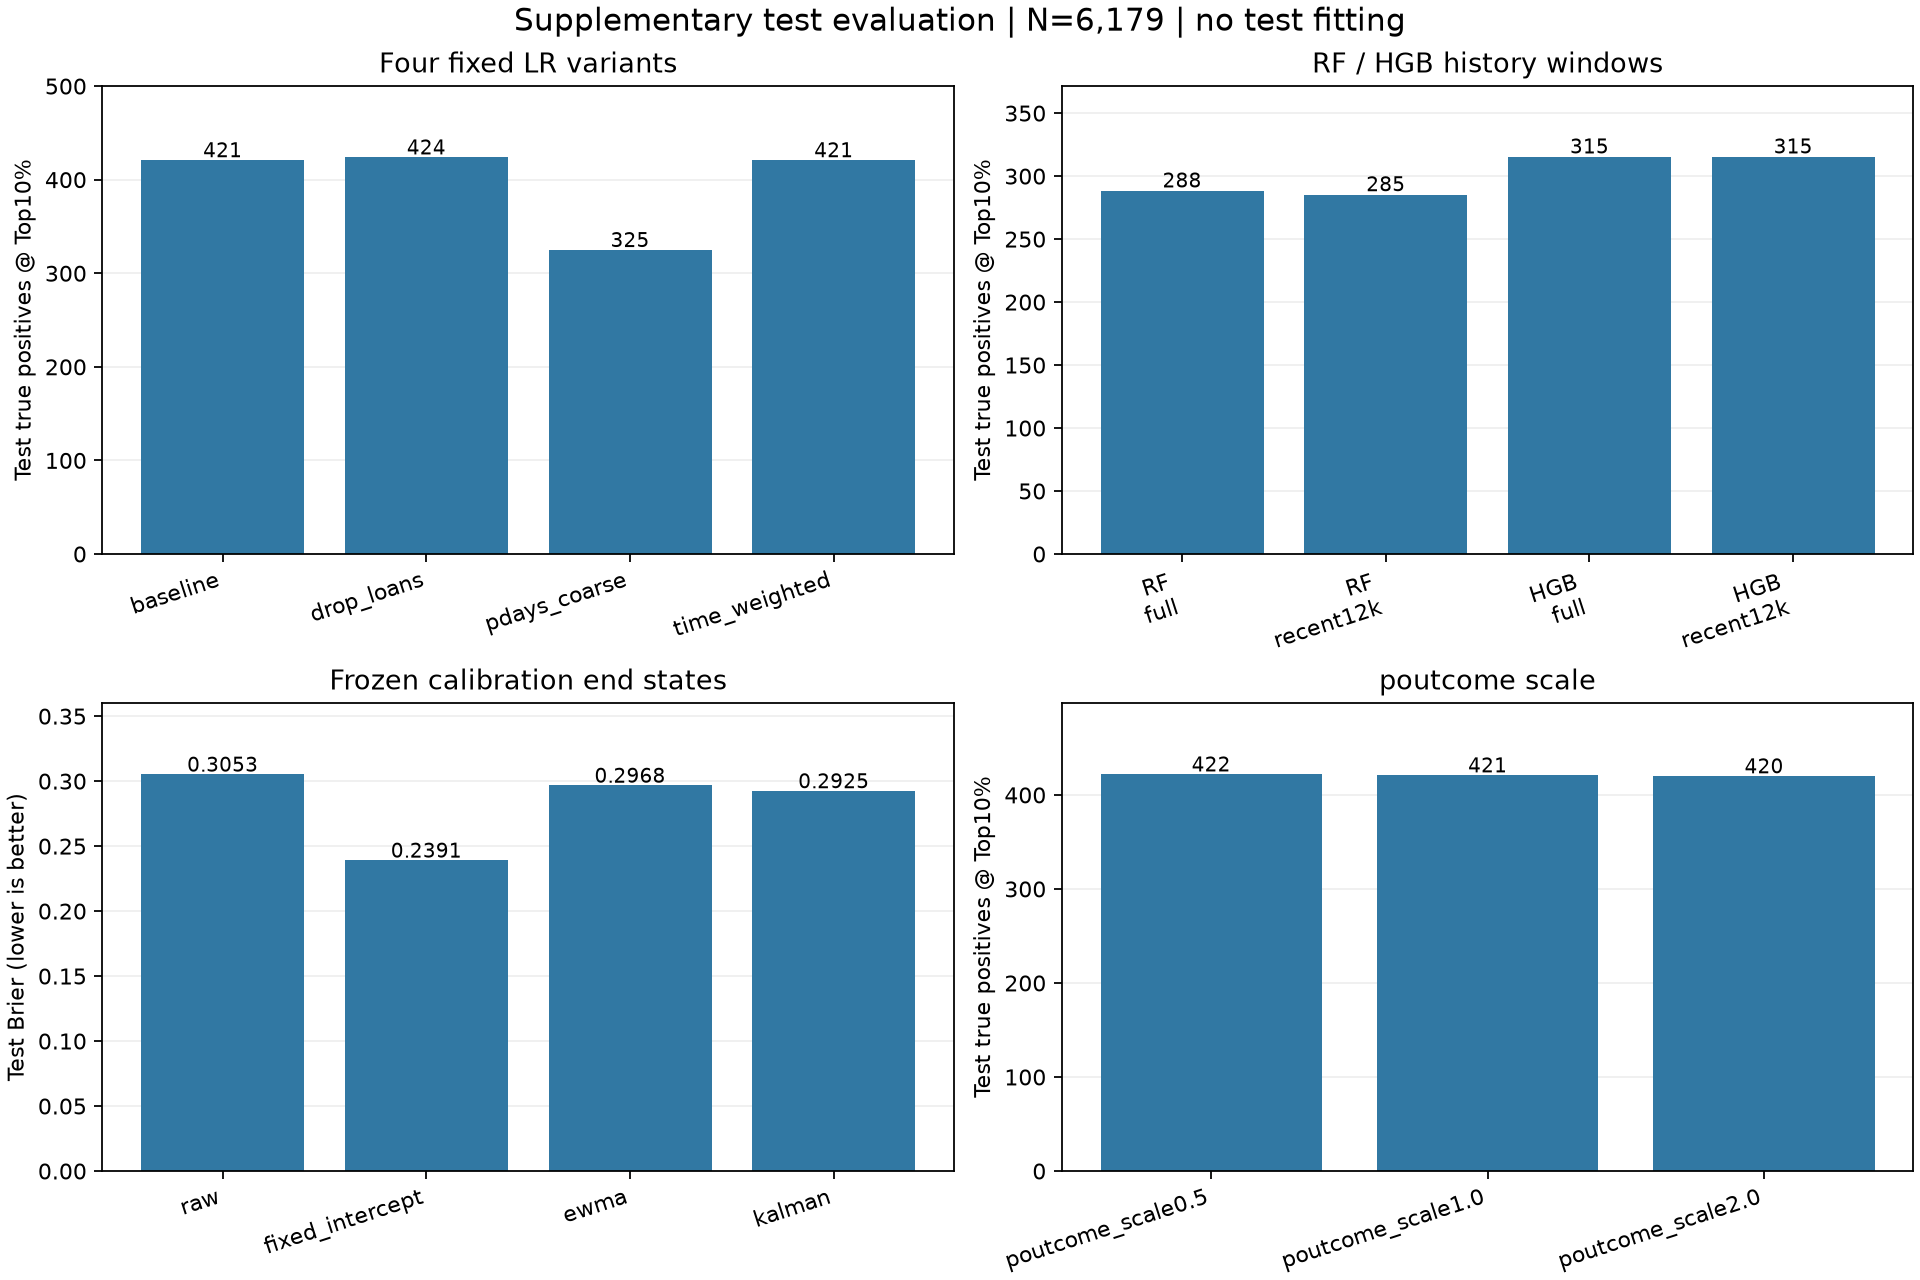


## 11. Discussion and conclusions / 结论与证据边界

**主作业与事后探索分开解释。** 第6节保留原首次冻结测试结果；
第7节起现在统一展示test，并把train/val开发依据作为补充。
本次407条分节引用中存在重复模型，不能把重复引用视为更多独立证据。

**联系LR参照。** 在相同test上，Top10联系618人、命中421，
Precision=68.1230%、Recall=17.7189%，
AUC=0.668025、AP=0.561969。
各支线必须与同信息范围、同预算的对照比较；不同范围模型不能仅凭名次解释某一字段的净贡献。

**最后四个单因素改动：**

- **drop_loans**：test Top10命中424（对照421，Δ=+3）；AUC 0.667793（Δ=-0.000232），AP 0.561859（Δ=-0.000110），Brier 0.305272（Δ=-0.000014）。
- **pdays_coarse**：test Top10命中325（对照421，Δ=-96）；AUC 0.593347（Δ=-0.074678），AP 0.465075（Δ=-0.096894），Brier 0.330592（Δ=+0.025306）。
- **time_weighted**：test Top10命中421（对照421，Δ=+0）；AUC 0.667372（Δ=-0.000653），AP 0.562519（Δ=+0.000550），Brier 0.302140（Δ=-0.003145）。

**训练窗口变短是否有效：**

- **RF**：最近12,000条相对全历史，test Top10命中 288→285，AUC 0.605081→0.566760，AP 0.462414→0.432624，Brier 0.298974→0.293116。
- **HGB**：最近12,000条相对全历史，test Top10命中 315→315，AUC 0.607053→0.574642，AP 0.489092→0.466255，Brier 0.295431→0.287013。

**动态校准终态迁移：**

- **fixed_intercept**：test Top10命中421（对照421，Δ=+0）；AUC 0.668025（Δ=+0.000000），AP 0.561969（Δ=+0.000000），Brier 0.239129（Δ=-0.066156）。
- **ewma**：test Top10命中421（对照421，Δ=+0）；AUC 0.668025（Δ=+0.000000），AP 0.561969（Δ=+0.000000），Brier 0.296768（Δ=-0.008517）。
- **kalman**：test Top10命中421（对照421，Δ=+0）；AUC 0.668025（Δ=+0.000000），AP 0.561969（Δ=+0.000000），Brier 0.292511（Δ=-0.012774）。

四种冻结截距保持test名单相同，差异主要体现在概率误差及固定0.5操作点。
W/E/S校准同样应看各自raw→校准后的Brier、log loss、ECE，而不能称为排序提升。
校准比较详见9.2的完整对照；不同基模型、校准窗口可能出现不同方向。

**可支持的结论范围。** train/val用于拟合、比较、校准与操作点冻结；本次test没有参与这些计算，
但它在更早阶段已经被查看，因此这些改动仍属于事后探索，独立泛化确认需要新的未来数据。
Top10命中变化、AP/AUC、Brier不必同方向，不能用单一指标宣布所有目标同时改善。
本次只补齐评价和展示，不依据test结果继续修改模型。

<details>
<summary>原版本总体结论（开发时期记录，当前判断以本节test解读为准）</summary>

## 11. Discussion and conclusions / 结论、局限与现实应用

**作业主结论。** 数据准备应由语义、训练分布与同模型对照共同检验。
共同unknown可放大关联；999与历史字段不能简单互换；高组内订购率不等于覆盖大量订购者；
标准化与删除列改变正则化几何，更多清理不必然提高预测能力。

**能力与边界。** 联系历史为已联系客户提供有限筛选价值，无法仅凭背景确定某人是否购买。
Precision、Recall、排序和概率质量回答不同问题；不平衡处理改变损失/概率尺度，不会创造新客户信息。
当前结果与信息不足、历史稀疏支持和跨期迁移共同存在相符，未量化三者各自因果贡献。

**严谨性限制。** 全量结构和test基础率曾被看过；后续方向是事后探索；val被反复使用；
相邻窗口共享训练历史、种子仅反映算法随机性。缺少日期、客户ID和标签成熟时间，不能证明真实时间/客户隔离。
Cramér’s V、系数及分组比例都是关联证据；没有营销随机对照，不能报告增量收益。
没有证明公平性满足任何标准：年龄、职业、学历可能影响名单，应监测分组选择率和错误，避免把群体关联当个体价值。

**面向现实的下一步。** 先补足客户ID、完整事件日期和预测时点可用的信息；采用带标签成熟间隔的滚动前向评估，
在过去窗口选择编码、校准和预算策略，最后在真正未见的未来批次确认。
监测基础率、分数与分组残差后再决定更新；近期加权和校准须另证，不应为了已知test比例强行调整。
业务若限制联系人数，固定预算比较Precision/Recall；有真实成本后再确定决策阈值，不能把F1当利润。

### Assignment alignment / 作业要求对应

| 教师要求 | 本草稿位置 |
|---|---|
| 数据画像、清理、转换及验证 | 1–4节 |
| 至少一个非显然问题与解释 | 共同缺失关联、历史字段语义、比例与覆盖、时间迁移 |
| 最少处理 vs 系统处理，同一种简单模型 | 4–6节，A/B/A_scaled及单因素对照 |
| 解释提升与退化，不以accuracy chasing为目标 | 5–10节保留失败结果与取舍 |
| 清晰代码、可重现流程和AI声明 | 可见Pipeline、CSV输入、已核验结果及本节声明 |
| ≤12分钟演示、成员贡献 | 小组自行完成，不能由本文件代替 |

### Contribution and AI declaration / 贡献与工具声明

| 成员姓名/学号 | 实际贡献 | 本人运行、理解和核对范围 |
|---|---|---|
| 待填写1 | 待填写 | 待确认 |
| 待填写2 | 待填写 | 待确认 |
| 待填写3 | 待填写 | 待确认 |
| 待填写4 | 待填写 | 待确认 |

工具使用草稿：Devin协助早期导入、EDA及准备决策；Codex协助代码、实验核查、图表与Notebook整理；
Grok提供审查建议。实际参与范围由小组确认。此次自动检查包括原件备份、核心拟合、历史数值复算和干净内核运行；
**不能代替成员对全部代码、理由和结论的理解与人工核对**，未预先声明所有成员已经完成。

依据：本地《Assignment Procedure.pdf》pp.1–3、5；数据说明来自UCI Bank Marketing原始字典；
课程Week1–4笔记用于数据准备、EDA和时间划分原则。
数据出处：[UCI数据记录](https://archive.ics.uci.edu/dataset/222/bank+marketing)、[DOI](https://doi.org/10.24432/C5K306)。

</details>


## Appendix A. Metrics and extended algorithms / 指标及扩展支线

| 指标 | 作用与解释 |
|---|---|
| Accuracy=(TP+TN)/N | 总体猜对比例；多数类占优时易掩盖低Recall |
| Precision=TP/(TP+FP) | 推荐名单里多少真订购；无人推荐时数学上未定义，统一结果表显示`—` |
| Recall=TP/(TP+FN) | 全部订购者找回多少 |
| F1=2PR/(P+R)=2TP/(2TP+FP+FN) | P为Precision，R为Recall；二者的调和平均，等价推导与零分母说明见第7节；不等于成本最优 |
| ROC-AUC | 随机正例得分高于随机负例的概率，平分计半；阈值不改变它 |
| AP | 按Recall增量加权的Precision；受基础率影响，不等同梯形PR-AUC |
| Brier / log loss | 概率质量，越低越好；log loss强惩罚自信错误，不含训练L2项 |
| Precision/Recall@K, lift | 固定预算下命中与覆盖；lift=Precision/该评价集基础率，不是增量收益 |
| ECE10 | 十等宽箱内预测均值与订购率偏差的加权均值；受分箱影响，不单独选模 |

**扩展算法边界：** 课程明确要求基本可解释模型。浅树属于该范围；RF、Balanced RF、HGB只作为已完成探索的附录记录，
不取代LR主实验，正式提交是否保留本附录应结合老师要求决定。
普通RF/加权RF/Balanced RF共用联系版信息和预处理；300棵树，min_samples_leaf=5，max_features=sqrt。
Balanced RF使用内部平衡抽样（all、replacement=True、bootstrap=False），与普通RF有多项机制差异。

### HGB扩展支线：test 完整性能

**主表全部为 test：6,179 人、2,376 个 yes（38.4528%）。** 共 8 个配置/参照，按 test ROC-AUC 降序展示前10项；排序仅用于阅读，不据此重新选择模型、阈值或窗口。所有阈值相关主表指标使用固定 Top10% 联系预算（618 人）；阈值数值列的“—”表示预算规则。

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|contact_HGB_d3_l210|test|top10|6179|2376|0.384528|—|0.101340|0.559404|0.435847|0.608351|0.464401|0.120791|0.191717|0.912963|0.516877|0.985502|0.316101|0.283188|618|1.207717|3472|331|2089|287|
|contact_HGB_d3_l21|test|top10|6179|2376|0.384528|—|0.104030|0.558575|0.431467|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.983940|0.314985|0.281086|618|1.203509|3471|332|2090|286|
|contact_HGB_d2_l21|test|top10|6179|2376|0.384528|—|0.099362|0.557952|0.431045|0.608675|0.466019|0.121212|0.192385|0.913226|0.517219|0.989178|0.317188|0.285166|618|1.211925|3473|330|2088|288|
|contact_HGB_d2_l210|test|top10|6179|2376|0.384528|—|0.095641|0.557651|0.429419|0.608027|0.462783|0.120370|0.191049|0.912700|0.516535|0.992648|0.318726|0.288887|618|1.203509|3471|332|2090|286|
|personal_HGB_d2_l210|test|top10|6179|2376|0.384528|—|0.087445|0.535779|0.416146|0.605761|0.451456|0.117424|0.186373|0.910860|0.514142|1.034281|0.324624|0.297083|618|1.174052|3464|339|2097|279|
|personal_HGB_d3_l210|test|top10|6179|2376|0.384528|—|0.092590|0.535308|0.419226|0.607380|0.459547|0.119529|0.189713|0.912175|0.515852|1.029071|0.322452|0.291938|618|1.195093|3469|334|2092|284|
|personal_HGB_d2_l21|test|top10|6179|2376|0.384528|—|0.092369|0.534359|0.416247|0.607056|0.457929|0.119108|0.189045|0.911912|0.515510|1.029460|0.322516|0.292159|618|1.190885|3468|335|2093|283|
|personal_HGB_d3_l21|test|top10|6179|2376|0.384528|—|0.096214|0.532719|0.418574|0.609322|0.469256|0.122054|0.193721|0.913752|0.517903|1.027655|0.321133|0.288314|618|1.220341|3475|328|2086|290|

<details>
<summary>固定0.5阈值：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_HGB_d2_l21|test|fixed_0.5|6179|2376|0.384528|0.500000|0.092369|0.534359|0.416247|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.029460|0.322516|0.292159|0|—|3803|0|2376|0|
|personal_HGB_d2_l210|test|fixed_0.5|6179|2376|0.384528|0.500000|0.087445|0.535779|0.416146|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.034281|0.324624|0.297083|0|—|3803|0|2376|0|
|personal_HGB_d3_l21|test|fixed_0.5|6179|2376|0.384528|0.500000|0.096214|0.532719|0.418574|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.027655|0.321133|0.288314|0|—|3803|0|2376|0|
|personal_HGB_d3_l210|test|fixed_0.5|6179|2376|0.384528|0.500000|0.092590|0.535308|0.419226|0.615472|—|0.000000|0.000000|1.000000|0.500000|1.029071|0.322452|0.291938|0|—|3803|0|2376|0|
|contact_HGB_d2_l21|test|fixed_0.5|6179|2376|0.384528|0.500000|0.099362|0.557952|0.431045|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.989178|0.317188|0.285166|0|—|3803|0|2376|0|
|contact_HGB_d2_l210|test|fixed_0.5|6179|2376|0.384528|0.500000|0.095641|0.557651|0.429419|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.992648|0.318726|0.288887|0|—|3803|0|2376|0|
|contact_HGB_d3_l21|test|fixed_0.5|6179|2376|0.384528|0.500000|0.104030|0.558575|0.431467|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.983940|0.314985|0.281086|0|—|3803|0|2376|0|
|contact_HGB_d3_l210|test|fixed_0.5|6179|2376|0.384528|0.500000|0.101340|0.559404|0.435847|0.615472|—|0.000000|0.000000|1.000000|0.500000|0.985502|0.316101|0.283188|0|—|3803|0|2376|0|

</details>

<details>
<summary>Top5%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_HGB_d2_l21|test|top5|6179|2376|0.384528|—|0.092369|0.534359|0.416247|0.611102|0.456311|0.059343|0.105028|0.955824|0.507584|1.029460|0.322516|0.292159|309|1.186677|3635|168|2235|141|
|personal_HGB_d2_l210|test|top5|6179|2376|0.384528|—|0.087445|0.535779|0.416146|0.610778|0.453074|0.058923|0.104283|0.955561|0.507242|1.034281|0.324624|0.297083|309|1.178260|3634|169|2236|140|
|personal_HGB_d3_l21|test|top5|6179|2376|0.384528|—|0.096214|0.532719|0.418574|0.613692|0.482201|0.062710|0.110987|0.957928|0.510319|1.027655|0.321133|0.288314|309|1.254006|3643|160|2227|149|
|personal_HGB_d3_l210|test|top5|6179|2376|0.384528|—|0.092590|0.535308|0.419226|0.612721|0.472492|0.061448|0.108752|0.957139|0.509293|1.029071|0.322452|0.291938|309|1.228757|3640|163|2230|146|
|contact_HGB_d2_l21|test|top5|6179|2376|0.384528|—|0.099362|0.557952|0.431045|0.612073|0.466019|0.060606|0.107263|0.956613|0.508610|0.989178|0.317188|0.285166|309|1.211925|3638|165|2232|144|
|contact_HGB_d2_l210|test|top5|6179|2376|0.384528|—|0.095641|0.557651|0.429419|0.610455|0.449838|0.058502|0.103538|0.955298|0.506900|0.992648|0.318726|0.288887|309|1.169844|3633|170|2237|139|
|contact_HGB_d3_l21|test|top5|6179|2376|0.384528|—|0.104030|0.558575|0.431467|0.618223|0.527508|0.068603|0.121415|0.961609|0.515106|0.983940|0.314985|0.281086|309|1.371832|3657|146|2213|163|
|contact_HGB_d3_l210|test|top5|6179|2376|0.384528|—|0.101340|0.559404|0.435847|0.618223|0.527508|0.068603|0.121415|0.961609|0.515106|0.985502|0.316101|0.283188|309|1.371832|3657|146|2213|163|

</details>

<details>
<summary>Top20%预算：全部 test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_HGB_d2_l21|test|top20|6179|2376|0.384528|—|0.092369|0.534359|0.416247|0.592167|0.441748|0.229798|0.302326|0.818564|0.524181|1.029460|0.322516|0.292159|1236|1.148804|3113|690|1830|546|
|personal_HGB_d2_l210|test|top20|6179|2376|0.384528|—|0.087445|0.535779|0.416146|0.595080|0.449029|0.233586|0.307309|0.820931|0.527258|1.034281|0.324624|0.297083|1236|1.167740|3122|681|1821|555|
|personal_HGB_d3_l21|test|top20|6179|2376|0.384528|—|0.096214|0.532719|0.418574|0.595727|0.450647|0.234428|0.308416|0.821457|0.527942|1.027655|0.321133|0.288314|1236|1.171948|3124|679|1819|557|
|personal_HGB_d3_l210|test|top20|6179|2376|0.384528|—|0.092590|0.535308|0.419226|0.596051|0.451456|0.234848|0.308970|0.821720|0.528284|1.029071|0.322452|0.291938|1236|1.174052|3125|678|1818|558|
|contact_HGB_d2_l21|test|top20|6179|2376|0.384528|—|0.099362|0.557952|0.431045|0.597346|0.454693|0.236532|0.311185|0.822771|0.529652|0.989178|0.317188|0.285166|1236|1.182469|3129|674|1814|562|
|contact_HGB_d2_l210|test|top20|6179|2376|0.384528|—|0.095641|0.557651|0.429419|0.598964|0.458738|0.238636|0.313953|0.824086|0.531361|0.992648|0.318726|0.288887|1236|1.192989|3134|669|1809|567|
|contact_HGB_d3_l21|test|top20|6179|2376|0.384528|—|0.104030|0.558575|0.431467|0.598964|0.458738|0.238636|0.313953|0.824086|0.531361|0.983940|0.314985|0.281086|1236|1.192989|3134|669|1809|567|
|contact_HGB_d3_l210|test|top20|6179|2376|0.384528|—|0.101340|0.559404|0.435847|0.596698|0.453074|0.235690|0.310078|0.822246|0.528968|0.985502|0.316101|0.283188|1236|1.178260|3127|676|1816|560|

</details>

<details>
<summary>仅用开发数据确定并冻结的阈值：test 指标</summary>

|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_HGB_d2_l21|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.169790|0.092369|0.534359|0.416247|0.602201|0.453409|0.167929|0.245086|0.873521|0.520725|1.029460|0.322516|0.292159|880|1.179131|3322|481|1977|399|
|personal_HGB_d2_l21|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.059577|0.092369|0.534359|0.416247|0.490371|0.397071|0.627525|0.486381|0.404681|0.516103|1.029460|0.322516|0.292159|3755|1.032617|1539|2264|885|1491|
|personal_HGB_d2_l21|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.169790|0.092369|0.534359|0.416247|0.602201|0.453409|0.167929|0.245086|0.873521|0.520725|1.029460|0.322516|0.292159|880|1.179131|3322|481|1977|399|
|personal_HGB_d2_l21|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.059577|0.092369|0.534359|0.416247|0.490371|0.397071|0.627525|0.486381|0.404681|0.516103|1.029460|0.322516|0.292159|3755|1.032617|1539|2264|885|1491|
|personal_HGB_d2_l210|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.088424|0.087445|0.535779|0.416146|0.593785|0.449925|0.253367|0.324179|0.806469|0.529918|1.034281|0.324624|0.297083|1338|1.170071|3067|736|1774|602|
|personal_HGB_d2_l210|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.056265|0.087445|0.535779|0.416146|0.473054|0.397004|0.713805|0.510229|0.322640|0.518222|1.034281|0.324624|0.297083|4272|1.032444|1227|2576|680|1696|
|personal_HGB_d2_l210|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.088424|0.087445|0.535779|0.416146|0.593785|0.449925|0.253367|0.324179|0.806469|0.529918|1.034281|0.324624|0.297083|1338|1.170071|3067|736|1774|602|
|personal_HGB_d2_l210|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.056265|0.087445|0.535779|0.416146|0.473054|0.397004|0.713805|0.510229|0.322640|0.518222|1.034281|0.324624|0.297083|4272|1.032444|1227|2576|680|1696|
|personal_HGB_d3_l21|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.099058|0.096214|0.532719|0.418574|0.591682|0.443764|0.244108|0.314961|0.808835|0.526471|1.027655|0.321133|0.288314|1307|1.154049|3076|727|1796|580|
|personal_HGB_d3_l21|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.325543|0.096214|0.532719|0.418574|0.614824|0.492537|0.055556|0.099849|0.964239|0.509897|1.027655|0.321133|0.288314|268|1.280887|3667|136|2244|132|
|personal_HGB_d3_l21|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.099058|0.096214|0.532719|0.418574|0.591682|0.443764|0.244108|0.314961|0.808835|0.526471|1.027655|0.321133|0.288314|1307|1.154049|3076|727|1796|580|
|personal_HGB_d3_l21|test|saved_dev_same_window_SELECTION_ONLY_0.325542737256|6179|2376|0.384528|0.325543|0.096214|0.532719|0.418574|0.614824|0.492537|0.055556|0.099849|0.964239|0.509897|1.027655|0.321133|0.288314|268|1.280887|3667|136|2244|132|
|personal_HGB_d3_l210|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.099626|0.092590|0.535308|0.419226|0.594595|0.450726|0.248316|0.320217|0.810939|0.529628|1.029071|0.322452|0.291938|1309|1.172153|3084|719|1786|590|
|personal_HGB_d3_l210|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.063264|0.092590|0.535308|0.419226|0.511571|0.401715|0.552189|0.465083|0.486195|0.519192|1.029071|0.322452|0.291938|3266|1.044695|1849|1954|1064|1312|
|personal_HGB_d3_l210|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.099626|0.092590|0.535308|0.419226|0.594595|0.450726|0.248316|0.320217|0.810939|0.529628|1.029071|0.322452|0.291938|1309|1.172153|3084|719|1786|590|
|personal_HGB_d3_l210|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.063264|0.092590|0.535308|0.419226|0.511571|0.401715|0.552189|0.465083|0.486195|0.519192|1.029071|0.322452|0.291938|3266|1.044695|1849|1954|1064|1312|
|contact_HGB_d2_l21|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.106210|0.099362|0.557952|0.431045|0.600097|0.460384|0.232323|0.308811|0.829871|0.531097|0.989178|0.317188|0.285166|1199|1.197269|3156|647|1824|552|
|contact_HGB_d2_l21|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.079726|0.099362|0.557952|0.431045|0.558505|0.427928|0.439815|0.433790|0.632658|0.536237|0.989178|0.317188|0.285166|2442|1.112865|2406|1397|1331|1045|
|contact_HGB_d2_l21|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.181407|0.099362|0.557952|0.431045|0.603981|0.454777|0.150253|0.225878|0.887457|0.518855|0.989178|0.317188|0.285166|785|1.182688|3375|428|2019|357|
|contact_HGB_d2_l21|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.106210|0.099362|0.557952|0.431045|0.600097|0.460384|0.232323|0.308811|0.829871|0.531097|0.989178|0.317188|0.285166|1199|1.197269|3156|647|1824|552|
|contact_HGB_d2_l21|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.079726|0.099362|0.557952|0.431045|0.558505|0.427928|0.439815|0.433790|0.632658|0.536237|0.989178|0.317188|0.285166|2442|1.112865|2406|1397|1331|1045|
|contact_HGB_d2_l21|test|saved_dev_same_window_SELECTION_ONLY_0.181407485984|6179|2376|0.384528|0.181407|0.099362|0.557952|0.431045|0.603981|0.454777|0.150253|0.225878|0.887457|0.518855|0.989178|0.317188|0.285166|785|1.182688|3375|428|2019|357|
|contact_HGB_d2_l210|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.117628|0.095641|0.557651|0.429419|0.603010|0.466019|0.222222|0.300940|0.840915|0.531569|0.992648|0.318726|0.288887|1133|1.211925|3198|605|1848|528|
|contact_HGB_d2_l210|test|saved_previous_window_TRANSFER_precision30|6179|2376|0.384528|0.075671|0.095641|0.557651|0.429419|0.541512|0.421612|0.517256|0.464562|0.556666|0.536961|0.992648|0.318726|0.288887|2915|1.096441|2117|1686|1147|1229|
|contact_HGB_d2_l210|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.164111|0.095641|0.557651|0.429419|0.604305|0.455598|0.148990|0.224548|0.888772|0.518881|0.992648|0.318726|0.288887|777|1.184824|3380|423|2022|354|
|contact_HGB_d2_l210|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.117628|0.095641|0.557651|0.429419|0.603010|0.466019|0.222222|0.300940|0.840915|0.531569|0.992648|0.318726|0.288887|1133|1.211925|3198|605|1848|528|
|contact_HGB_d2_l210|test|saved_dev_previous_window_TRANSFER|6179|2376|0.384528|0.075671|0.095641|0.557651|0.429419|0.541512|0.421612|0.517256|0.464562|0.556666|0.536961|0.992648|0.318726|0.288887|2915|1.096441|2117|1686|1147|1229|
|contact_HGB_d2_l210|test|saved_dev_same_window_SELECTION_ONLY_0.164110518074|6179|2376|0.384528|0.164111|0.095641|0.557651|0.429419|0.604305|0.455598|0.148990|0.224548|0.888772|0.518881|0.992648|0.318726|0.288887|777|1.184824|3380|423|2022|354|
|contact_HGB_d3_l21|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.115241|0.104030|0.558575|0.431467|0.595404|0.454810|0.262626|0.332978|0.803313|0.532970|0.983940|0.314985|0.281086|1372|1.182775|3055|748|1752|624|
|contact_HGB_d3_l21|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.209300|0.104030|0.558575|0.431467|0.608513|0.465041|0.120370|0.191240|0.913489|0.516930|0.983940|0.314985|0.281086|615|1.209380|3474|329|2090|286|
|contact_HGB_d3_l21|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.115241|0.104030|0.558575|0.431467|0.595404|0.454810|0.262626|0.332978|0.803313|0.532970|0.983940|0.314985|0.281086|1372|1.182775|3055|748|1752|624|
|contact_HGB_d3_l21|test|saved_dev_same_window_SELECTION_ONLY_0.209300037797|6179|2376|0.384528|0.209300|0.104030|0.558575|0.431467|0.608513|0.465041|0.120370|0.191240|0.913489|0.516930|0.983940|0.314985|0.281086|615|1.209380|3474|329|2090|286|
|contact_HGB_d3_l210|test|saved_same_window_SELECTION_ONLY_precision30|6179|2376|0.384528|0.110984|0.101340|0.559404|0.435847|0.593785|0.452415|0.268098|0.336681|0.797265|0.532681|0.985502|0.316101|0.283188|1408|1.176545|3032|771|1739|637|
|contact_HGB_d3_l210|test|saved_same_window_SELECTION_ONLY_precision40|6179|2376|0.384528|0.171507|0.101340|0.559404|0.435847|0.605761|0.461440|0.151094|0.227647|0.889824|0.520459|0.985502|0.316101|0.283188|778|1.200015|3384|419|2017|359|
|contact_HGB_d3_l210|test|saved_dev_same_window_SELECTION_ONLY|6179|2376|0.384528|0.110984|0.101340|0.559404|0.435847|0.593785|0.452415|0.268098|0.336681|0.797265|0.532681|0.985502|0.316101|0.283188|1408|1.176545|3032|771|1739|637|
|contact_HGB_d3_l210|test|saved_dev_same_window_SELECTION_ONLY_0.171506816083|6179|2376|0.384528|0.171507|0.101340|0.559404|0.435847|0.605761|0.461440|0.151094|0.227647|0.889824|0.520459|0.985502|0.316101|0.283188|778|1.200015|3384|419|2017|359|

</details>

<details>
<summary>train/val 拟合、调参与 test 来源</summary>

|Model|训练与开发依据|预测来源键|
|---|---|---|
|personal_HGB_d2_l21|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|boosting_error_audit__personal_HGB_d2_l21|
|personal_HGB_d2_l210|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|boosting_error_audit__personal_HGB_d2_l210|
|personal_HGB_d3_l21|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|boosting_error_audit__personal_HGB_d3_l21|
|personal_HGB_d3_l210|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|boosting_error_audit__personal_HGB_d3_l210|
|contact_HGB_d2_l21|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|boosting_error_audit__contact_HGB_d2_l21|
|contact_HGB_d2_l210|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|boosting_error_audit__contact_HGB_d2_l210|
|contact_HGB_d3_l21|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|boosting_error_audit__contact_HGB_d3_l21|
|contact_HGB_d3_l210|原 train 拟合；前向开发窗口/val 选配置和阈值；复用历史 test 预测|boosting_error_audit__contact_HGB_d3_l210|

</details>

<details>
<summary>按 poutcome 切片：test 完整指标（先用全体规则确定名单，再切组）</summary>

|poutcome|Model|Split|Rule|N|Yes|Yes rate|Threshold|Mean p|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Specificity|Balanced Acc|Log loss|Brier|ECE10|Contacts|Lift|TN|FP|FN|TP|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|failure|personal_HGB_d2_l21|test|fixed_0.5|1492|443|0.296917|0.500000|0.093599|0.524132|0.312300|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.824084|0.253756|0.207064|0|—|1049|0|443|0|
|nonexistent|personal_HGB_d2_l21|test|fixed_0.5|3516|1113|0.316553|0.500000|0.089678|0.533688|0.346680|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.868512|0.268366|0.226875|0|—|2403|0|1113|0|
|success|personal_HGB_d2_l21|test|fixed_0.5|1171|820|0.700256|0.500000|0.098881|0.519646|0.725149|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.774391|0.572717|0.601375|0|—|351|0|820|0|
|failure|personal_HGB_d2_l21|test|top5|1492|443|0.296917|—|0.093599|0.524132|0.312300|0.682976|0.302632|0.051919|0.088632|0.949476|0.500697|0.824084|0.253756|0.207064|76|1.019247|996|53|420|23|
|nonexistent|personal_HGB_d2_l21|test|top5|3516|1113|0.316553|—|0.089678|0.533688|0.346680|0.673777|0.397590|0.059299|0.103206|0.958385|0.508842|0.868512|0.268366|0.226875|166|1.256000|2303|100|1047|66|
|success|personal_HGB_d2_l21|test|top5|1171|820|0.700256|—|0.098881|0.519646|0.725149|0.331341|0.776119|0.063415|0.117249|0.957265|0.510340|1.774391|0.572717|0.601375|67|1.108336|336|15|768|52|
|failure|personal_HGB_d2_l21|test|top10|1492|443|0.296917|—|0.093599|0.524132|0.312300|0.663539|0.309677|0.108352|0.160535|0.897998|0.503175|0.824084|0.253756|0.207064|155|1.042977|942|107|395|48|
|nonexistent|personal_HGB_d2_l21|test|top10|3516|1113|0.316553|—|0.089678|0.533688|0.346680|0.664960|0.402985|0.121294|0.186464|0.916771|0.519032|0.868512|0.268366|0.226875|335|1.273042|2203|200|978|135|
|success|personal_HGB_d2_l21|test|top10|1171|820|0.700256|—|0.098881|0.519646|0.725149|0.361230|0.781250|0.121951|0.210970|0.920228|0.521090|1.774391|0.572717|0.601375|128|1.115663|323|28|720|100|
|failure|personal_HGB_d2_l21|test|top20|1492|443|0.296917|—|0.093599|0.524132|0.312300|0.634048|0.335463|0.237020|0.277778|0.801716|0.519368|0.824084|0.253756|0.207064|313|1.129822|841|208|338|105|
|nonexistent|personal_HGB_d2_l21|test|top20|3516|1113|0.316553|—|0.089678|0.533688|0.346680|0.633675|0.362205|0.206649|0.263158|0.831461|0.519055|0.868512|0.268366|0.226875|635|1.144215|1998|405|883|230|
|success|personal_HGB_d2_l21|test|top20|1171|820|0.700256|—|0.098881|0.519646|0.725149|0.414176|0.732639|0.257317|0.380866|0.780627|0.518972|1.774391|0.572717|0.601375|288|1.046244|274|77|609|211|
|failure|personal_HGB_d2_l210|test|fixed_0.5|1492|443|0.296917|0.500000|0.088505|0.526987|0.311605|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.824543|0.254359|0.208412|0|—|1049|0|443|0|
|nonexistent|personal_HGB_d2_l210|test|fixed_0.5|3516|1113|0.316553|0.500000|0.085100|0.533963|0.345169|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.871764|0.269826|0.231453|0|—|2403|0|1113|0|
|success|personal_HGB_d2_l210|test|fixed_0.5|1171|820|0.700256|0.500000|0.093135|0.520869|0.728137|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.789482|0.578686|0.607121|0|—|351|0|820|0|
|failure|personal_HGB_d2_l210|test|top5|1492|443|0.296917|—|0.088505|0.526987|0.311605|0.681635|0.277778|0.045147|0.077670|0.950429|0.497788|0.824543|0.254359|0.208412|72|0.935541|997|52|423|20|
|nonexistent|personal_HGB_d2_l210|test|top5|3516|1113|0.316553|—|0.085100|0.533963|0.345169|0.672639|0.388235|0.059299|0.102884|0.956721|0.508010|0.871764|0.269826|0.231453|170|1.226447|2299|104|1047|66|
|success|personal_HGB_d2_l210|test|top5|1171|820|0.700256|—|0.093135|0.520869|0.728137|0.334757|0.805970|0.065854|0.121759|0.962963|0.514408|1.789482|0.578686|0.607121|67|1.150965|338|13|766|54|
|failure|personal_HGB_d2_l210|test|top10|1492|443|0.296917|—|0.088505|0.526987|0.311605|0.662198|0.308176|0.110609|0.162791|0.895138|0.502874|0.824543|0.254359|0.208412|159|1.037920|939|110|394|49|
|nonexistent|personal_HGB_d2_l210|test|top10|3516|1113|0.316553|—|0.085100|0.533963|0.345169|0.664107|0.398204|0.119497|0.183829|0.916355|0.517926|0.871764|0.269826|0.231453|334|1.257937|2202|201|980|133|
|success|personal_HGB_d2_l210|test|top10|1171|820|0.700256|—|0.093135|0.520869|0.728137|0.358668|0.776000|0.118293|0.205291|0.920228|0.519260|1.789482|0.578686|0.607121|125|1.108166|323|28|723|97|
|failure|personal_HGB_d2_l210|test|top20|1492|443|0.296917|—|0.088505|0.526987|0.311605|0.635389|0.338658|0.239278|0.280423|0.802669|0.520973|0.824543|0.254359|0.208412|313|1.140582|842|207|337|106|
|nonexistent|personal_HGB_d2_l210|test|top20|3516|1113|0.316553|—|0.085100|0.533963|0.345169|0.637372|0.372240|0.212040|0.270177|0.834374|0.523207|0.871764|0.269826|0.231453|634|1.175916|2005|398|877|236|
|success|personal_HGB_d2_l210|test|top20|1171|820|0.700256|—|0.093135|0.520869|0.728137|0.416738|0.737024|0.259756|0.384130|0.783476|0.521616|1.789482|0.578686|0.607121|289|1.052507|275|76|607|213|
|failure|personal_HGB_d3_l21|test|fixed_0.5|1492|443|0.296917|0.500000|0.097355|0.522854|0.311901|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.824995|0.253699|0.207867|0|—|1049|0|443|0|
|nonexistent|personal_HGB_d3_l21|test|fixed_0.5|3516|1113|0.316553|0.500000|0.093308|0.532321|0.350845|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.867606|0.267383|0.223244|0|—|2403|0|1113|0|
|success|personal_HGB_d3_l21|test|fixed_0.5|1171|820|0.700256|0.500000|0.103484|0.519448|0.722631|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.766426|0.568443|0.596773|0|—|351|0|820|0|
|failure|personal_HGB_d3_l21|test|top5|1492|443|0.296917|—|0.097355|0.522854|0.311901|0.682306|0.287671|0.047404|0.081395|0.950429|0.498917|0.824995|0.253699|0.207867|73|0.968861|997|52|422|21|
|nonexistent|personal_HGB_d3_l21|test|top5|3516|1113|0.316553|—|0.093308|0.532321|0.350845|0.676337|0.424242|0.062893|0.109546|0.960466|0.511680|0.867606|0.267383|0.223244|165|1.340194|2308|95|1043|70|
|success|personal_HGB_d3_l21|test|top5|1171|820|0.700256|—|0.103484|0.519448|0.722631|0.338173|0.816901|0.070732|0.130191|0.962963|0.516847|1.766426|0.568443|0.596773|71|1.166575|338|13|762|58|
|failure|personal_HGB_d3_l21|test|top10|1492|443|0.296917|—|0.097355|0.522854|0.311901|0.662198|0.308176|0.110609|0.162791|0.895138|0.502874|0.824995|0.253699|0.207867|159|1.037920|939|110|394|49|
|nonexistent|personal_HGB_d3_l21|test|top10|3516|1113|0.316553|—|0.093308|0.532321|0.350845|0.668373|0.418462|0.122192|0.189152|0.921348|0.521770|0.867606|0.267383|0.223244|325|1.321932|2214|189|977|136|
|success|personal_HGB_d3_l21|test|top10|1171|820|0.700256|—|0.103484|0.519448|0.722631|0.364646|0.783582|0.128049|0.220126|0.917379|0.522714|1.766426|0.568443|0.596773|134|1.118993|322|29|715|105|
|failure|personal_HGB_d3_l21|test|top20|1492|443|0.296917|—|0.097355|0.522854|0.311901|0.634718|0.337580|0.239278|0.280053|0.801716|0.520497|0.824995|0.253699|0.207867|314|1.136950|841|208|337|106|
|nonexistent|personal_HGB_d3_l21|test|top20|3516|1113|0.316553|—|0.093308|0.532321|0.350845|0.637656|0.372425|0.211141|0.269495|0.835206|0.523174|0.867606|0.267383|0.223244|631|1.176501|2007|396|878|235|
|success|personal_HGB_d3_l21|test|top20|1171|820|0.700256|—|0.103484|0.519448|0.722631|0.420154|0.742268|0.263415|0.388839|0.786325|0.524870|1.766426|0.568443|0.596773|291|1.059995|276|75|604|216|
|failure|personal_HGB_d3_l210|test|fixed_0.5|1492|443|0.296917|0.500000|0.093645|0.525305|0.312823|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.824754|0.254116|0.204530|0|—|1049|0|443|0|
|nonexistent|personal_HGB_d3_l210|test|fixed_0.5|3516|1113|0.316553|0.500000|0.089996|0.534305|0.351345|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.867631|0.268136|0.226557|0|—|2403|0|1113|0|
|success|personal_HGB_d3_l210|test|fixed_0.5|1171|820|0.700256|0.500000|0.099036|0.521880|0.723116|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.774130|0.572607|0.601220|0|—|351|0|820|0|
|failure|personal_HGB_d3_l210|test|top5|1492|443|0.296917|—|0.093645|0.525305|0.312823|0.681635|0.277778|0.045147|0.077670|0.950429|0.497788|0.824754|0.254116|0.204530|72|0.935541|997|52|423|20|
|nonexistent|personal_HGB_d3_l210|test|top5|3516|1113|0.316553|—|0.089996|0.534305|0.351345|0.676906|0.432749|0.066487|0.115265|0.959634|0.513060|0.867631|0.268136|0.226557|171|1.367065|2306|97|1039|74|
|success|personal_HGB_d3_l210|test|top5|1171|820|0.700256|—|0.099036|0.521880|0.723116|0.332195|0.787879|0.063415|0.117381|0.960114|0.511764|1.774130|0.572607|0.601220|66|1.125129|337|14|768|52|
|failure|personal_HGB_d3_l210|test|top10|1492|443|0.296917|—|0.093645|0.525305|0.312823|0.663539|0.309677|0.108352|0.160535|0.897998|0.503175|0.824754|0.254116|0.204530|155|1.042977|942|107|395|48|
|nonexistent|personal_HGB_d3_l210|test|top10|3516|1113|0.316553|—|0.089996|0.534305|0.351345|0.665245|0.404192|0.121294|0.186593|0.917187|0.519240|0.867631|0.268136|0.226557|334|1.276853|2204|199|978|135|
|success|personal_HGB_d3_l210|test|top10|1171|820|0.700256|—|0.099036|0.521880|0.723116|0.362084|0.782946|0.123171|0.212856|0.920228|0.521699|1.774130|0.572607|0.601220|129|1.118085|323|28|719|101|
|failure|personal_HGB_d3_l210|test|top20|1492|443|0.296917|—|0.093645|0.525305|0.312823|0.632708|0.334385|0.239278|0.278947|0.798856|0.519067|0.824754|0.254116|0.204530|317|1.126190|838|211|337|106|
|nonexistent|personal_HGB_d3_l210|test|top20|3516|1113|0.316553|—|0.089996|0.534305|0.351345|0.638510|0.374204|0.211141|0.269960|0.836454|0.523798|0.867631|0.268136|0.226557|628|1.182121|2010|393|878|235|
|success|personal_HGB_d3_l210|test|top20|1171|820|0.700256|—|0.099036|0.521880|0.723116|0.421862|0.745704|0.264634|0.390639|0.789174|0.526904|1.774130|0.572607|0.601220|291|1.064902|277|74|603|217|
|failure|contact_HGB_d2_l21|test|fixed_0.5|1492|443|0.296917|0.500000|0.101338|0.531391|0.317532|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.792392|0.249144|0.199663|0|—|1049|0|443|0|
|nonexistent|contact_HGB_d2_l21|test|fixed_0.5|3516|1113|0.316553|0.500000|0.095343|0.560395|0.357363|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.839222|0.264858|0.222359|0|—|2403|0|1113|0|
|success|contact_HGB_d2_l21|test|fixed_0.5|1171|820|0.700256|0.500000|0.108914|0.522829|0.725383|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.690158|0.561009|0.591342|0|—|351|0|820|0|
|failure|contact_HGB_d2_l21|test|top5|1492|443|0.296917|—|0.101338|0.531391|0.317532|0.686327|0.244898|0.027088|0.048780|0.964728|0.495908|0.792392|0.249144|0.199663|49|0.824803|1012|37|431|12|
|nonexistent|contact_HGB_d2_l21|test|top5|3516|1113|0.316553|—|0.095343|0.560395|0.357363|0.674915|0.420213|0.070979|0.121445|0.954640|0.512810|0.839222|0.264858|0.222359|188|1.327465|2294|109|1034|79|
|success|contact_HGB_d2_l21|test|top5|1171|820|0.700256|—|0.108914|0.522829|0.725383|0.328779|0.736111|0.064634|0.118834|0.945869|0.505252|1.690158|0.561009|0.591342|72|1.051203|332|19|767|53|
|failure|contact_HGB_d2_l21|test|top10|1492|443|0.296917|—|0.101338|0.531391|0.317532|0.670912|0.355422|0.133183|0.193760|0.897998|0.515590|0.792392|0.249144|0.199663|166|1.197041|942|107|384|59|
|nonexistent|contact_HGB_d2_l21|test|top10|3516|1113|0.316553|—|0.095343|0.560395|0.357363|0.662969|0.381579|0.104223|0.163726|0.921764|0.512994|0.839222|0.264858|0.222359|304|1.205419|2215|188|997|116|
|success|contact_HGB_d2_l21|test|top10|1171|820|0.700256|—|0.108914|0.522829|0.725383|0.366354|0.763514|0.137805|0.233471|0.900285|0.519045|1.690158|0.561009|0.591342|148|1.090335|316|35|707|113|
|failure|contact_HGB_d2_l21|test|top20|1492|443|0.296917|—|0.101338|0.531391|0.317532|0.635389|0.339683|0.241535|0.282322|0.801716|0.521625|0.792392|0.249144|0.199663|315|1.144032|841|208|336|107|
|nonexistent|contact_HGB_d2_l21|test|top20|3516|1113|0.316553|—|0.095343|0.560395|0.357363|0.638225|0.371567|0.206649|0.265589|0.838119|0.522384|0.839222|0.264858|0.222359|619|1.173791|2014|389|883|230|
|success|contact_HGB_d2_l21|test|top20|1171|820|0.700256|—|0.108914|0.522829|0.725383|0.426132|0.745033|0.274390|0.401070|0.780627|0.527509|1.690158|0.561009|0.591342|302|1.063944|274|77|595|225|
|failure|contact_HGB_d2_l210|test|fixed_0.5|1492|443|0.296917|0.500000|0.098596|0.534143|0.320465|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.790329|0.249307|0.198320|0|—|1049|0|443|0|
|nonexistent|contact_HGB_d2_l210|test|fixed_0.5|3516|1113|0.316553|0.500000|0.091725|0.562831|0.359670|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.841276|0.265716|0.224828|0|—|2403|0|1113|0|
|success|contact_HGB_d2_l210|test|fixed_0.5|1171|820|0.700256|0.500000|0.103635|0.524081|0.726592|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.704933|0.566342|0.596621|0|—|351|0|820|0|
|failure|contact_HGB_d2_l210|test|top5|1492|443|0.296917|—|0.098596|0.534143|0.320465|0.682976|0.312500|0.056433|0.095602|0.947569|0.502001|0.790329|0.249307|0.198320|80|1.052483|994|55|418|25|
|nonexistent|contact_HGB_d2_l210|test|top5|3516|1113|0.316553|—|0.091725|0.562831|0.359670|0.674346|0.404762|0.061096|0.106167|0.958385|0.509741|0.841276|0.265716|0.224828|168|1.278655|2303|100|1045|68|
|success|contact_HGB_d2_l210|test|top5|1171|820|0.700256|—|0.103635|0.524081|0.726592|0.326217|0.754098|0.056098|0.104427|0.957265|0.506681|1.704933|0.566342|0.596621|61|1.076889|336|15|774|46|
|failure|contact_HGB_d2_l210|test|top10|1492|443|0.296917|—|0.098596|0.534143|0.320465|0.670241|0.351515|0.130926|0.190789|0.897998|0.514462|0.790329|0.249307|0.198320|165|1.183884|942|107|385|58|
|nonexistent|contact_HGB_d2_l210|test|top10|3516|1113|0.316553|—|0.091725|0.562831|0.359670|0.663254|0.383607|0.105121|0.165021|0.921764|0.513443|0.841276|0.265716|0.224828|305|1.211824|2215|188|996|117|
|success|contact_HGB_d2_l210|test|top10|1171|820|0.700256|—|0.103635|0.524081|0.726592|0.362938|0.750000|0.135366|0.229339|0.894587|0.514976|1.704933|0.566342|0.596621|148|1.071037|314|37|709|111|
|failure|contact_HGB_d2_l210|test|top20|1492|443|0.296917|—|0.098596|0.534143|0.320465|0.632708|0.336449|0.243792|0.282723|0.796949|0.520371|0.790329|0.249307|0.198320|321|1.133141|836|213|335|108|
|nonexistent|contact_HGB_d2_l210|test|top20|3516|1113|0.316553|—|0.091725|0.562831|0.359670|0.641354|0.379479|0.209344|0.269832|0.841448|0.525396|0.841276|0.265716|0.224828|614|1.198785|2022|381|880|233|
|success|contact_HGB_d2_l210|test|top20|1171|820|0.700256|—|0.103635|0.524081|0.726592|0.428693|0.750831|0.275610|0.403211|0.786325|0.530967|1.704933|0.566342|0.596621|301|1.072223|276|75|594|226|
|failure|contact_HGB_d3_l21|test|fixed_0.5|1492|443|0.296917|0.500000|0.101874|0.529233|0.315044|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.802138|0.250056|0.202177|0|—|1049|0|443|0|
|nonexistent|contact_HGB_d3_l21|test|fixed_0.5|3516|1113|0.316553|0.500000|0.100840|0.557100|0.359065|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.833659|0.263025|0.216289|0|—|2403|0|1113|0|
|success|contact_HGB_d3_l21|test|fixed_0.5|1171|820|0.700256|0.500000|0.116354|0.521833|0.717717|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.666808|0.553729|0.584588|0|—|351|0|820|0|
|failure|contact_HGB_d3_l21|test|top5|1492|443|0.296917|—|0.101874|0.529233|0.315044|0.697721|0.100000|0.002257|0.004415|0.991420|0.496839|0.802138|0.250056|0.202177|10|0.336795|1040|9|442|1|
|nonexistent|contact_HGB_d3_l21|test|top5|3516|1113|0.316553|—|0.100840|0.557100|0.359065|0.676906|0.444976|0.083558|0.140696|0.951727|0.517642|0.833659|0.263025|0.216289|209|1.405693|2287|116|1020|93|
|success|contact_HGB_d3_l21|test|top5|1171|820|0.700256|—|0.116354|0.521833|0.717717|0.340734|0.766667|0.084146|0.151648|0.940171|0.512159|1.666808|0.553729|0.584588|90|1.094837|330|21|751|69|
|failure|contact_HGB_d3_l21|test|top10|1492|443|0.296917|—|0.101874|0.529233|0.315044|0.672922|0.346939|0.115124|0.172881|0.908484|0.511804|0.802138|0.250056|0.202177|147|1.168471|953|96|392|51|
|nonexistent|contact_HGB_d3_l21|test|top10|3516|1113|0.316553|—|0.100840|0.557100|0.359065|0.660694|0.374214|0.106918|0.166317|0.917187|0.512053|0.833659|0.263025|0.216289|318|1.182153|2204|199|994|119|
|success|contact_HGB_d3_l21|test|top10|1171|820|0.700256|—|0.116354|0.521833|0.717717|0.367208|0.758170|0.141463|0.238438|0.894587|0.518025|1.666808|0.553729|0.584588|153|1.082704|314|37|704|116|
|failure|contact_HGB_d3_l21|test|top20|1492|443|0.296917|—|0.101874|0.529233|0.315044|0.636729|0.340836|0.239278|0.281167|0.804576|0.521927|0.802138|0.250056|0.202177|311|1.147917|844|205|337|106|
|nonexistent|contact_HGB_d3_l21|test|top20|3516|1113|0.316553|—|0.100840|0.557100|0.359065|0.641923|0.381877|0.212040|0.272675|0.841032|0.526536|0.833659|0.263025|0.216289|618|1.206361|2021|382|877|236|
|success|contact_HGB_d3_l21|test|top20|1171|820|0.700256|—|0.116354|0.521833|0.717717|0.421862|0.732899|0.274390|0.399290|0.766382|0.520386|1.666808|0.553729|0.584588|307|1.046616|269|82|595|225|
|failure|contact_HGB_d3_l210|test|fixed_0.5|1492|443|0.296917|0.500000|0.101061|0.532481|0.318616|0.703083|—|0.000000|0.000000|1.000000|0.500000|0.795692|0.249491|0.195855|0|—|1049|0|443|0|
|nonexistent|contact_HGB_d3_l210|test|fixed_0.5|3516|1113|0.316553|0.500000|0.097921|0.559369|0.361042|0.683447|—|0.000000|0.000000|1.000000|0.500000|0.835225|0.263836|0.219963|0|—|2403|0|1113|0|
|success|contact_HGB_d3_l210|test|fixed_0.5|1171|820|0.700256|0.500000|0.111961|0.524234|0.724839|0.299744|—|0.000000|0.000000|1.000000|0.500000|1.678560|0.557899|0.588295|0|—|351|0|820|0|
|failure|contact_HGB_d3_l210|test|top5|1492|443|0.296917|—|0.101061|0.532481|0.318616|0.698391|0.230769|0.006772|0.013158|0.990467|0.498620|0.795692|0.249491|0.195855|13|0.777218|1039|10|440|3|
|nonexistent|contact_HGB_d3_l210|test|top5|3516|1113|0.316553|—|0.097921|0.559369|0.361042|0.676621|0.442857|0.083558|0.140590|0.951311|0.517434|0.835225|0.263836|0.219963|210|1.398999|2286|117|1020|93|
|success|contact_HGB_d3_l210|test|top5|1171|820|0.700256|—|0.111961|0.524234|0.724839|0.340734|0.779070|0.081707|0.147903|0.945869|0.513788|1.678560|0.557899|0.588295|86|1.112550|332|19|753|67|
|failure|contact_HGB_d3_l210|test|top10|1492|443|0.296917|—|0.101061|0.532481|0.318616|0.672922|0.348993|0.117381|0.175676|0.907531|0.512456|0.795692|0.249491|0.195855|149|1.175390|952|97|391|52|
|nonexistent|contact_HGB_d3_l210|test|top10|3516|1113|0.316553|—|0.097921|0.559369|0.361042|0.661263|0.376582|0.106918|0.166550|0.918019|0.512469|0.835225|0.263836|0.219963|316|1.189635|2206|197|994|119|
|success|contact_HGB_d3_l210|test|top10|1171|820|0.700256|—|0.111961|0.524234|0.724839|0.367208|0.758170|0.141463|0.238438|0.894587|0.518025|1.678560|0.557899|0.588295|153|1.082704|314|37|704|116|
|failure|contact_HGB_d3_l210|test|top20|1492|443|0.296917|—|0.101061|0.532481|0.318616|0.634718|0.336538|0.237020|0.278146|0.802669|0.519845|0.795692|0.249491|0.195855|312|1.133443|842|207|338|105|
|nonexistent|contact_HGB_d3_l210|test|top20|3516|1113|0.316553|—|0.097921|0.559369|0.361042|0.638794|0.373997|0.209344|0.268433|0.837703|0.523523|0.835225|0.263836|0.219963|623|1.181467|2013|390|880|233|
|success|contact_HGB_d3_l210|test|top20|1171|820|0.700256|—|0.111961|0.524234|0.724839|0.421862|0.737542|0.270732|0.396075|0.774929|0.522830|1.678560|0.557899|0.588295|301|1.053245|272|79|598|222|

</details>

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### HGB扩展支线：完整性能

下表为每个模型在val的Top10%口径；全部0.5口径、其他窗口和原有阈值规则见展开表。数值由本地保存预测重新计算。

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_HGB_d2_l21|val|top10|6178|0.1065|—|0.5907|0.1691|0.8378|0.2217|0.2082|0.2147|0.3468|0.0956|137|481|521|5039|
|personal_HGB_d2_l210|val|top10|6178|0.1065|—|0.5953|0.1721|0.8391|0.2282|0.2143|0.2210|0.3466|0.0957|141|477|517|5043|
|personal_HGB_d3_l21|val|top10|6178|0.1065|—|0.5916|0.1701|0.8398|0.2314|0.2173|0.2241|0.3469|0.0956|143|475|515|5045|
|personal_HGB_d3_l210|val|top10|6178|0.1065|—|0.5936|0.1711|0.8401|0.2330|0.2188|0.2257|0.3467|0.0956|144|474|514|5046|
|contact_HGB_d2_l21|val|top10|6178|0.1065|—|0.5906|0.1773|0.8375|0.2201|0.2067|0.2132|0.3387|0.0945|136|482|522|5038|
|contact_HGB_d2_l210|val|top10|6178|0.1065|—|0.5889|0.1711|0.8375|0.2201|0.2067|0.2132|0.3391|0.0947|136|482|522|5038|
|contact_HGB_d3_l21|val|top10|6178|0.1065|—|0.5954|0.1778|0.8394|0.2298|0.2158|0.2226|0.3380|0.0943|142|476|516|5044|
|contact_HGB_d3_l210|val|top10|6178|0.1065|—|0.5936|0.1761|0.8388|0.2265|0.2128|0.2194|0.3381|0.0944|140|478|518|5042|

<details>
<summary>展开全部窗口、种子、0.5及原阈值指标（95行）</summary>

|Model|Window|Rule|N|Yes rate|Threshold|ROC-AUC|AP|Accuracy|Precision|Recall|F1|Log loss|Brier|TP|FP|FN|TN|
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
|personal_HGB_d2_l21|D1|fixed_0.5|4000|0.0655|0.5|0.5146|0.0703|0.9345|—|0.0000|0.0000|0.2526|0.0621|0|0|262|3738|
|personal_HGB_d2_l21|D1|top10|4000|0.0655|—|0.5146|0.0703|0.8510|0.0825|0.1260|0.0997|0.2526|0.0621|33|367|229|3371|
|personal_HGB_d2_l210|D1|fixed_0.5|4000|0.0655|0.5|0.5091|0.0679|0.9345|—|0.0000|0.0000|0.2523|0.0621|0|0|262|3738|
|personal_HGB_d2_l210|D1|top10|4000|0.0655|—|0.5091|0.0679|0.8485|0.0700|0.1069|0.0846|0.2523|0.0621|28|372|234|3366|
|personal_HGB_d3_l21|D1|fixed_0.5|4000|0.0655|0.5|0.5129|0.0697|0.9345|—|0.0000|0.0000|0.2539|0.0621|0|0|262|3738|
|personal_HGB_d3_l21|D1|top10|4000|0.0655|—|0.5129|0.0697|0.8520|0.0875|0.1336|0.1057|0.2539|0.0621|35|365|227|3373|
|personal_HGB_d3_l210|D1|fixed_0.5|4000|0.0655|0.5|0.5023|0.0669|0.9345|—|0.0000|0.0000|0.2534|0.0621|0|0|262|3738|
|personal_HGB_d3_l210|D1|top10|4000|0.0655|—|0.5023|0.0669|0.8485|0.0700|0.1069|0.0846|0.2534|0.0621|28|372|234|3366|
|contact_HGB_d2_l21|D1|fixed_0.5|4000|0.0655|0.5|0.5204|0.0706|0.9345|—|0.0000|0.0000|0.2520|0.0620|0|0|262|3738|
|contact_HGB_d2_l21|D1|top10|4000|0.0655|—|0.5204|0.0706|0.8510|0.0825|0.1260|0.0997|0.2520|0.0620|33|367|229|3371|
|contact_HGB_d2_l210|D1|fixed_0.5|4000|0.0655|0.5|0.5129|0.0671|0.9345|—|0.0000|0.0000|0.2522|0.0621|0|0|262|3738|
|contact_HGB_d2_l210|D1|top10|4000|0.0655|—|0.5129|0.0671|0.8470|0.0625|0.0954|0.0755|0.2522|0.0621|25|375|237|3363|
|contact_HGB_d3_l21|D1|fixed_0.5|4000|0.0655|0.5|0.5199|0.0704|0.9345|—|0.0000|0.0000|0.2531|0.0621|0|0|262|3738|
|contact_HGB_d3_l21|D1|top10|4000|0.0655|—|0.5199|0.0704|0.8510|0.0825|0.1260|0.0997|0.2531|0.0621|33|367|229|3371|
|contact_HGB_d3_l210|D1|fixed_0.5|4000|0.0655|0.5|0.5157|0.0691|0.9345|—|0.0000|0.0000|0.2526|0.0621|0|0|262|3738|
|contact_HGB_d3_l210|D1|top10|4000|0.0655|—|0.5157|0.0691|0.8505|0.0800|0.1221|0.0967|0.2526|0.0621|32|368|230|3370|
|personal_HGB_d2_l21|D2|fixed_0.5|4000|0.0580|0.5|0.5071|0.0606|0.9420|—|0.0000|0.0000|0.2256|0.0550|0|0|232|3768|
|personal_HGB_d2_l21|D2|top10|4000|0.0580|—|0.5071|0.0606|0.8550|0.0650|0.1121|0.0823|0.2256|0.0550|26|374|206|3394|
|personal_HGB_d2_l210|D2|fixed_0.5|4000|0.0580|0.5|0.5058|0.0601|0.9420|—|0.0000|0.0000|0.2252|0.0549|0|0|232|3768|
|personal_HGB_d2_l210|D2|top10|4000|0.0580|—|0.5058|0.0601|0.8555|0.0675|0.1164|0.0854|0.2252|0.0549|27|373|205|3395|
|personal_HGB_d3_l21|D2|fixed_0.5|4000|0.0580|0.5|0.5048|0.0597|0.9420|—|0.0000|0.0000|0.2263|0.0550|0|0|232|3768|
|personal_HGB_d3_l21|D2|top10|4000|0.0580|—|0.5048|0.0597|0.8535|0.0575|0.0991|0.0728|0.2263|0.0550|23|377|209|3391|
|personal_HGB_d3_l210|D2|fixed_0.5|4000|0.0580|0.5|0.4947|0.0582|0.9420|—|0.0000|0.0000|0.2259|0.0550|0|0|232|3768|
|personal_HGB_d3_l210|D2|top10|4000|0.0580|—|0.4947|0.0582|0.8540|0.0600|0.1034|0.0759|0.2259|0.0550|24|376|208|3392|
|contact_HGB_d2_l21|D2|fixed_0.5|4000|0.0580|0.5|0.5259|0.0643|0.9420|—|0.0000|0.0000|0.2224|0.0548|0|0|232|3768|
|contact_HGB_d2_l21|D2|top10|4000|0.0580|—|0.5259|0.0643|0.8535|0.0575|0.0991|0.0728|0.2224|0.0548|23|377|209|3391|
|contact_HGB_d2_l210|D2|fixed_0.5|4000|0.0580|0.5|0.5240|0.0629|0.9420|—|0.0000|0.0000|0.2225|0.0548|0|0|232|3768|
|contact_HGB_d2_l210|D2|top10|4000|0.0580|—|0.5240|0.0629|0.8530|0.0550|0.0948|0.0696|0.2225|0.0548|22|378|210|3390|
|contact_HGB_d3_l21|D2|fixed_0.5|4000|0.0580|0.5|0.5069|0.0586|0.9420|—|0.0000|0.0000|0.2252|0.0551|0|0|232|3768|
|contact_HGB_d3_l21|D2|top10|4000|0.0580|—|0.5069|0.0586|0.8520|0.0500|0.0862|0.0633|0.2252|0.0551|20|380|212|3388|
|contact_HGB_d3_l210|D2|fixed_0.5|4000|0.0580|0.5|0.5057|0.0591|0.9420|—|0.0000|0.0000|0.2241|0.0550|0|0|232|3768|
|contact_HGB_d3_l210|D2|top10|4000|0.0580|—|0.5057|0.0591|0.8500|0.0400|0.0690|0.0506|0.2241|0.0550|16|384|216|3384|
|personal_HGB_d2_l21|D3|fixed_0.5|4000|0.0485|0.5|0.4706|0.0462|0.9515|—|0.0000|0.0000|0.1960|0.0463|0|0|194|3806|
|personal_HGB_d2_l21|D3|top10|4000|0.0485|—|0.4706|0.0462|0.8590|0.0375|0.0773|0.0505|0.1960|0.0463|15|385|179|3421|
|personal_HGB_d2_l210|D3|fixed_0.5|4000|0.0485|0.5|0.4742|0.0451|0.9515|—|0.0000|0.0000|0.1957|0.0463|0|0|194|3806|
|personal_HGB_d2_l210|D3|top10|4000|0.0485|—|0.4742|0.0451|0.8585|0.0350|0.0722|0.0471|0.1957|0.0463|14|386|180|3420|
|personal_HGB_d3_l21|D3|fixed_0.5|4000|0.0485|0.5|0.4518|0.0453|0.9515|—|0.0000|0.0000|0.1975|0.0464|0|0|194|3806|
|personal_HGB_d3_l21|D3|top10|4000|0.0485|—|0.4518|0.0453|0.8595|0.0400|0.0825|0.0539|0.1975|0.0464|16|384|178|3422|
|personal_HGB_d3_l210|D3|fixed_0.5|4000|0.0485|0.5|0.4652|0.0462|0.9515|—|0.0000|0.0000|0.1962|0.0463|0|0|194|3806|
|personal_HGB_d3_l210|D3|top10|4000|0.0485|—|0.4652|0.0462|0.8600|0.0425|0.0876|0.0572|0.1962|0.0463|17|383|177|3423|
|contact_HGB_d2_l21|D3|fixed_0.5|4000|0.0485|0.5|0.4907|0.0473|0.9515|—|0.0000|0.0000|0.1976|0.0466|0|0|194|3806|
|contact_HGB_d2_l21|D3|top10|4000|0.0485|—|0.4907|0.0473|0.8590|0.0375|0.0773|0.0505|0.1976|0.0466|15|385|179|3421|
|contact_HGB_d2_l210|D3|fixed_0.5|4000|0.0485|0.5|0.4911|0.0472|0.9515|—|0.0000|0.0000|0.1974|0.0465|0|0|194|3806|
|contact_HGB_d2_l210|D3|top10|4000|0.0485|—|0.4911|0.0472|0.8600|0.0425|0.0876|0.0572|0.1974|0.0465|17|383|177|3423|
|contact_HGB_d3_l21|D3|fixed_0.5|4000|0.0485|0.5|0.4908|0.0483|0.9515|—|0.0000|0.0000|0.1983|0.0467|0|0|194|3806|
|contact_HGB_d3_l21|D3|top10|4000|0.0485|—|0.4908|0.0483|0.8590|0.0375|0.0773|0.0505|0.1983|0.0467|15|385|179|3421|
|contact_HGB_d3_l210|D3|fixed_0.5|4000|0.0485|0.5|0.4975|0.0476|0.9515|—|0.0000|0.0000|0.1978|0.0466|0|0|194|3806|
|contact_HGB_d3_l210|D3|top10|4000|0.0485|—|0.4975|0.0476|0.8605|0.0450|0.0928|0.0606|0.1978|0.0466|18|382|176|3424|
|personal_HGB_d2_l21|D4|fixed_0.5|4831|0.1031|0.5|0.6080|0.1648|0.8969|—|0.0000|0.0000|0.3545|0.0952|0|0|498|4333|
|personal_HGB_d2_l21|D4|top10|4831|0.1031|—|0.6080|0.1648|0.8352|0.1921|0.1867|0.1894|0.3545|0.0952|93|391|405|3942|
|personal_HGB_d2_l210|D4|fixed_0.5|4831|0.1031|0.5|0.6268|0.1778|0.8969|—|0.0000|0.0000|0.3547|0.0952|0|0|498|4333|
|personal_HGB_d2_l210|D4|top10|4831|0.1031|—|0.6268|0.1778|0.8377|0.2045|0.1988|0.2016|0.3547|0.0952|99|385|399|3948|
|personal_HGB_d3_l21|D4|fixed_0.5|4831|0.1031|0.5|0.5627|0.1302|0.8969|—|0.0000|0.0000|0.3563|0.0953|0|0|498|4333|
|personal_HGB_d3_l21|D4|top10|4831|0.1031|—|0.5627|0.1302|0.8249|0.1405|0.1365|0.1385|0.3563|0.0953|68|416|430|3917|
|personal_HGB_d3_l210|D4|fixed_0.5|4831|0.1031|0.5|0.5875|0.1488|0.8969|—|0.0000|0.0000|0.3549|0.0952|0|0|498|4333|
|personal_HGB_d3_l210|D4|top10|4831|0.1031|—|0.5875|0.1488|0.8319|0.1756|0.1707|0.1731|0.3549|0.0952|85|399|413|3934|
|contact_HGB_d2_l21|D4|fixed_0.5|4831|0.1031|0.5|0.4994|0.1223|0.8969|—|0.0000|0.0000|0.3520|0.0948|0|0|498|4333|
|contact_HGB_d2_l21|D4|top10|4831|0.1031|—|0.4994|0.1223|0.8203|0.1178|0.1145|0.1161|0.3520|0.0948|57|427|441|3906|
|contact_HGB_d2_l210|D4|fixed_0.5|4831|0.1031|0.5|0.4910|0.1173|0.8969|—|0.0000|0.0000|0.3525|0.0949|0|0|498|4333|
|contact_HGB_d2_l210|D4|top10|4831|0.1031|—|0.4910|0.1173|0.8187|0.1095|0.1064|0.1079|0.3525|0.0949|53|431|445|3902|
|contact_HGB_d3_l21|D4|fixed_0.5|4831|0.1031|0.5|0.4764|0.1067|0.8969|—|0.0000|0.0000|0.3537|0.0949|0|0|498|4333|
|contact_HGB_d3_l21|D4|top10|4831|0.1031|—|0.4764|0.1067|0.8191|0.1116|0.1084|0.1100|0.3537|0.0949|54|430|444|3903|
|contact_HGB_d3_l210|D4|fixed_0.5|4831|0.1031|0.5|0.4952|0.1084|0.8969|—|0.0000|0.0000|0.3524|0.0948|0|0|498|4333|
|contact_HGB_d3_l210|D4|top10|4831|0.1031|—|0.4952|0.1084|0.8207|0.1198|0.1165|0.1181|0.3524|0.0948|58|426|440|3907|
|personal_HGB_d2_l21|val|fixed_0.5|6178|0.1065|0.5|0.5907|0.1691|0.8935|—|0.0000|0.0000|0.3468|0.0956|0|0|658|5520|
|personal_HGB_d2_l210|val|fixed_0.5|6178|0.1065|0.5|0.5953|0.1721|0.8935|—|0.0000|0.0000|0.3466|0.0957|0|0|658|5520|
|personal_HGB_d3_l21|val|fixed_0.5|6178|0.1065|0.5|0.5916|0.1701|0.8935|—|0.0000|0.0000|0.3469|0.0956|0|0|658|5520|
|personal_HGB_d3_l210|val|fixed_0.5|6178|0.1065|0.5|0.5936|0.1711|0.8935|—|0.0000|0.0000|0.3467|0.0956|0|0|658|5520|
|contact_HGB_d2_l21|val|fixed_0.5|6178|0.1065|0.5|0.5906|0.1773|0.8935|—|0.0000|0.0000|0.3387|0.0945|0|0|658|5520|
|contact_HGB_d2_l210|val|fixed_0.5|6178|0.1065|0.5|0.5889|0.1711|0.8935|—|0.0000|0.0000|0.3391|0.0947|0|0|658|5520|
|contact_HGB_d3_l21|val|fixed_0.5|6178|0.1065|0.5|0.5954|0.1778|0.8935|—|0.0000|0.0000|0.3380|0.0943|0|0|658|5520|
|contact_HGB_d3_l210|val|fixed_0.5|6178|0.1065|0.5|0.5936|0.1761|0.8935|—|0.0000|0.0000|0.3381|0.0944|0|0|658|5520|
|personal_HGB_d2_l21|D4|same_window_SELECTION_ONLY|4831|0.1031|0.059577412|0.6080|0.1648|0.8868|0.3377|0.1024|0.1572|0.3545|0.0952|51|100|447|4233|
|personal_HGB_d2_l210|D4|same_window_SELECTION_ONLY|4831|0.1031|0.056264821|0.6268|0.1778|0.8849|0.3294|0.1124|0.1677|0.3547|0.0952|56|114|442|4219|
|personal_HGB_d3_l210|D4|same_window_SELECTION_ONLY|4831|0.1031|0.063264487|0.5875|0.1488|0.8884|0.3010|0.0622|0.1032|0.3549|0.0952|31|72|467|4261|
|contact_HGB_d2_l21|D4|same_window_SELECTION_ONLY|4831|0.1031|0.079726265|0.4994|0.1223|0.8953|0.3667|0.0221|0.0417|0.3520|0.0948|11|19|487|4314|
|contact_HGB_d2_l210|D4|same_window_SELECTION_ONLY|4831|0.1031|0.075670849|0.4910|0.1173|0.8944|0.3125|0.0201|0.0377|0.3525|0.0949|10|22|488|4311|
|personal_HGB_d2_l21|val|same_window_SELECTION_ONLY|6178|0.1065|0.16979007|0.5907|0.1691|0.8849|0.3037|0.0623|0.1034|0.3468|0.0956|41|94|617|5426|
|personal_HGB_d2_l21|val|previous_window_TRANSFER|6178|0.1065|0.059577412|0.5907|0.1691|0.5704|0.1279|0.5213|0.2054|0.3468|0.0956|343|2339|315|3181|
|personal_HGB_d2_l210|val|same_window_SELECTION_ONLY|6178|0.1065|0.08842444|0.5953|0.1721|0.8762|0.3026|0.1246|0.1765|0.3466|0.0957|82|189|576|5331|
|personal_HGB_d2_l210|val|previous_window_TRANSFER|6178|0.1065|0.056264821|0.5953|0.1721|0.5283|0.1277|0.5881|0.2099|0.3466|0.0957|387|2643|271|2877|
|personal_HGB_d3_l21|val|same_window_SELECTION_ONLY|6178|0.1065|0.099058156|0.5916|0.1701|0.8773|0.3000|0.1140|0.1652|0.3469|0.0956|75|175|583|5345|
|personal_HGB_d3_l21|val|same_window_SELECTION_ONLY|6178|0.1065|0.32554274|0.5916|0.1701|0.8925|0.4062|0.0198|0.0377|0.3469|0.0956|13|19|645|5501|
|personal_HGB_d3_l210|val|same_window_SELECTION_ONLY|6178|0.1065|0.099625881|0.5936|0.1711|0.8780|0.3049|0.1140|0.1659|0.3467|0.0956|75|171|583|5349|
|personal_HGB_d3_l210|val|previous_window_TRANSFER|6178|0.1065|0.063264487|0.5936|0.1711|0.6894|0.1464|0.3967|0.2138|0.3467|0.0956|261|1522|397|3998|
|contact_HGB_d2_l21|val|same_window_SELECTION_ONLY|6178|0.1065|0.10620952|0.5906|0.1773|0.8789|0.3009|0.1033|0.1538|0.3387|0.0945|68|158|590|5362|
|contact_HGB_d2_l21|val|previous_window_TRANSFER|6178|0.1065|0.079726265|0.5906|0.1773|0.7781|0.1774|0.2979|0.2223|0.3387|0.0945|196|909|462|4611|
|contact_HGB_d2_l21|val|same_window_SELECTION_ONLY|6178|0.1065|0.18140749|0.5906|0.1773|0.8903|0.4074|0.0669|0.1149|0.3387|0.0945|44|64|614|5456|
|contact_HGB_d2_l210|val|same_window_SELECTION_ONLY|6178|0.1065|0.11762788|0.5889|0.1711|0.8815|0.3221|0.1018|0.1547|0.3391|0.0947|67|141|591|5379|
|contact_HGB_d2_l210|val|previous_window_TRANSFER|6178|0.1065|0.075670849|0.5889|0.1711|0.7120|0.1486|0.3602|0.2104|0.3391|0.0947|237|1358|421|4162|
|contact_HGB_d2_l210|val|same_window_SELECTION_ONLY|6178|0.1065|0.16411052|0.5889|0.1711|0.8904|0.4112|0.0669|0.1150|0.3391|0.0947|44|63|614|5457|
|contact_HGB_d3_l21|val|same_window_SELECTION_ONLY|6178|0.1065|0.11524085|0.5954|0.1778|0.8754|0.3056|0.1337|0.1860|0.3380|0.0943|88|200|570|5320|
|contact_HGB_d3_l21|val|same_window_SELECTION_ONLY|6178|0.1065|0.20930004|0.5954|0.1778|0.8912|0.4079|0.0471|0.0845|0.3380|0.0943|31|45|627|5475|
|contact_HGB_d3_l210|val|same_window_SELECTION_ONLY|6178|0.1065|0.11098352|0.5936|0.1761|0.8734|0.3000|0.1413|0.1921|0.3381|0.0944|93|217|565|5303|
|contact_HGB_d3_l210|val|same_window_SELECTION_ONLY|6178|0.1065|0.17150682|0.5936|0.1761|0.8904|0.4112|0.0669|0.1150|0.3381|0.0944|44|63|614|5457|

</details>


</details>


RF、加权RF、BRF的事后test指标见9.1；HGB各扩展配置的test完整结果见上表。
窗口RF/HGB的配对test差异见10.1。种子范围只是重复运行差异，不是泛化置信区间。

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

RF支线未超过同信息范围联系LR的val Top10表现；BRF相对普通RF的三个种子变化为+6、−3、+4个命中，
不能称稳定改进。HGB在该受控范围内也未解决区分瓶颈。种子范围不是泛化置信区间。

## Appendix B. Optional atlas and evidence access / 可选全字段图与来源

可选图直接从当前CSV的train/val计算，不读取历史结果文件。年龄按5岁，计数按语义分组；连续宏观字段按train四分位点分组，并显式覆盖超出训练范围的值。
下方开关默认关闭以保持文件清爽；打开后重画每个字段的train/val组内比例与val组人数。
连续宏观值按train规则显示，age按5岁；duration仅为事后描述、不能进入模型。

</details>


**复现边界。** 本文件保留原核心/联系模型的代码与执行顺序，默认重新拟合8个核心/联系模型。
第7节起的补充test结果以表格和图保存在本文件中；各节也保留实际训练范围、开发阶段选择依据与原train/val结果。
Run All不会重新训练全部扩展模型、搜索参数或新增补充test预测。
精简仓库不包含扩展实验的模型、逐样本预测和完整重训工具，不能将阅读这些嵌入结果等同于从头复现全部实验。

本次test展示更新已完成指标复算、结构及部分渲染检查，尚未对更新后的整本Notebook重新执行Run All。

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

**复现边界。** 本文件默认重新拟合8个核心/联系模型；扩展实验使用本地已完成预测重新核对后写入正文的结果表。
运行全部不重新搜索或重训数百个历史模型，正文表格也不会被新结果静默覆盖。精简仓库只提供原始CSV和本文件内的核心分析代码；扩展实验的完整重训工具不随仓库发布。

历史test已被多次查看；此处的测试表不能称为新的独立盲测。开发阶段各次试错仍按原协议区分，失败结果不删除。


</details>


### 完整指标如何解读

主表Split一律为test。所有候选给出ROC-AUC、AP、Accuracy、Precision、Recall、F1、
Specificity、Balanced Accuracy、log loss、Brier、ECE10、TN/FP/FN/TP、联系人数与Lift；
Top5/10/20及固定0.5分别报告，存在已保存开发阈值时也全部保留。
组内指标是在全体test名单确定后切片；不是对每个poutcome组重新选Top10。
Precision无定义时显示“—”，不能擅自填0掩盖无预测正例的情况。
test正类率与val不同，不能只比较二者的AP/Precision绝对值来判断模型改进。

<details>
<summary>原 train/val 开发结果与选择依据（历史原文，不是当前 test 主结果）</summary>

### 完整指标如何解读

所有候选都补齐ROC-AUC、AP、Accuracy、Precision、Recall、F1、log loss、Brier和TN/FP/FN/TP。
Top10表可直接比较同一个窗口、同样联系人数下“找到多少人、误报多少人”；0.5表说明固定默认阈值的行为；原F1/Precision规则说明历史实际选择的取舍。
模型之间不能只凭Accuracy判断优劣，更不能跨不同基础率的窗口把Precision差异全归因于模型改进。


</details>


## Appendix C. Development code / train与val过程补充

**以下代码及其原保存输出用于复现train拟合、val比较、系数和开发图表，不是test主结果。**
代码顺序与原Notebook一致；没有为展示test而重新运行这些拟合。
第7–10节及扩展算法正文中的静态表才是统一的事后test评价。



In [11]:
"""Train-only fitted representations for exploratory personal/macro comparisons."""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

MACRO=['emp.var.rate','cons.price.idx','cons.conf.idx','euribor3m','nr.employed']
PERSONAL=['job','marital','education','default','housing','loan']

class HistoryFeatures(TransformerMixin,BaseEstimator):
    def fit(self,X,y=None):
        assert 'y' not in X and 'duration' not in X
        self.feature_names_in_=np.asarray(X.columns,dtype=object)
        return self
    def transform(self,X):
        assert 'y' not in X and 'duration' not in X
        z=X.copy()
        z['campaign_log']=np.log1p(z.campaign)
        z['previous_group']=np.where(z.previous==0,'0',np.where(z.previous==1,'1','2plus'))
        z['pdays_known']=(z.pdays!=999).astype(float)
        z['pdays_log']=np.where(z.pdays!=999,np.log1p(z.pdays),0.)
        return z

def build_contact_representation(spec):
    drop=set(spec.get('drop',[]))
    cat=[c for c in PERSONAL+['contact','month','day_of_week','poutcome'] if c not in drop]
    if spec['history']>=1 and 'previous' not in drop: cat+=['previous_group']
    num=['campaign_log'] if 'campaign' not in drop else []
    # Binary indicator intentionally unscaled; rare indicator is not upweighted.
    binary=['pdays_known'] if spec['history']>=2 and 'pdays' not in drop else []
    if spec['history']>=3 and 'pdays' not in drop: num+=['pdays_log']
    groups=[('cat',OneHotEncoder(handle_unknown='ignore',drop=None),cat)]
    if num: groups.append(('num',StandardScaler(),num))
    if binary: groups.append(('binary','passthrough',binary))
    if 'age' not in drop:
        age=StandardScaler() if spec['age']=='linear' else SplineTransformer(n_knots=4,degree=2,knots='quantile',extrapolation='constant',include_bias=False)
        groups.append(('age',age,['age']))
    if spec.get('macro_penalty'):
        groups.append(('macro',StandardScaler(),MACRO))
    weights={'macro':1/np.sqrt(spec['macro_penalty'])} if spec.get('macro_penalty') else None
    pre=ColumnTransformer(groups,transformer_weights=weights,sparse_threshold=1.0)
    penalty_options={'l1_ratio':0.0} if tuple(int(v) for v in sklearn.__version__.split('.')[:2])>=(1,8) else {'penalty':'l2'}
    clf=LogisticRegression(C=1,solver='lbfgs',tol=1e-7,max_iter=20000,class_weight=None,**penalty_options)
    return Pipeline([('features',HistoryFeatures()),('preprocess',pre),('classifier',clf)])

budget,n_contact,N,positive_rate,ROC-AUC,AP,Accuracy,Precision,Recall,F1,Log loss,Brier,TP,FP,FN,TN,lift
0.0500,309,6178,0.1065,0.6593,0.2147,0.8801,0.3657,0.1717,0.2337,0.3354,0.0943,113,196,545,5324,3.4335
0.1000,618,6178,0.1065,0.6593,0.2147,0.8491,0.2783,0.2614,0.2696,0.3354,0.0943,172,446,486,5074,2.6131
0.2000,1236,6178,0.1065,0.6593,0.2147,0.7747,0.2031,0.3815,0.2650,0.3354,0.0943,251,985,407,4535,1.9067


model,rule,threshold,ROC-AUC,AP,Accuracy,Precision,Recall,F1,Log loss,Brier,tp,fp,fn,tn
contact_LR_spline_C0.01,fixed_0.5,0.5000,0.6593,0.2147,0.8935,—,0.0000,0.0000,0.3354,0.0943,0,0,658,5520
contact_LR_spline_C0.01,val_F1_selection_only,0.0873,0.6593,0.2147,0.8592,0.3037,0.2492,0.2738,0.3354,0.0943,164,376,494,5144


Contact LR val AUC/AP: 0.659345 0.214682


poutcome,n,yes,observed,predicted
failure,1808,106,0.0586,0.0620
nonexistent,4218,485,0.1150,0.0685
success,152,67,0.4408,0.1815


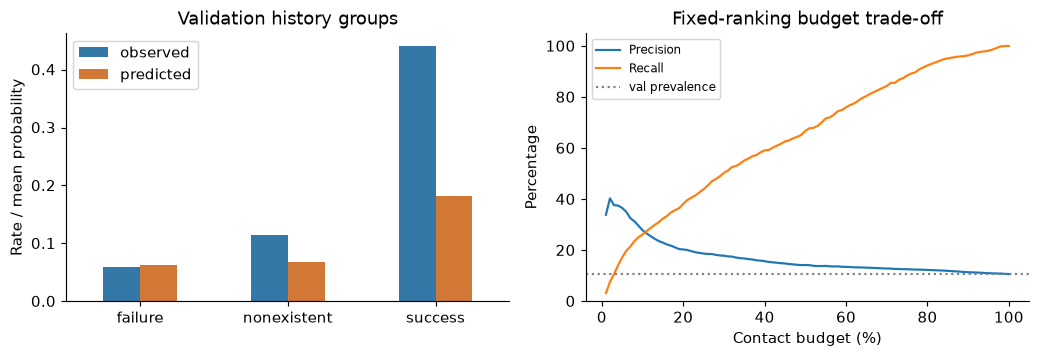

In [12]:
contact_spec={'age':'spline','history':3,'macro_penalty':None,'drop':['month','day_of_week']}
contact_model=None
contact_model=build_contact_representation(contact_spec)
contact_model.set_params(classifier__C=.01)
with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always');contact_model.fit(X_train,y_train)
assert contact_model.named_steps['classifier'].n_iter_[0]<20000
assert not any(issubclass(w.category,ConvergenceWarning) for w in caught)
rerun_contact=contact_model.predict_proba(X_val)[:,1]
contact_p=rerun_contact

def budget_metrics(y,p,fraction):
    y=np.asarray(y);p=np.asarray(p)
    k=int(np.ceil(len(y)*fraction))
    order=np.lexsort((np.arange(len(p)), -p))[:k]  # Original row-order tie break; no labels.
    tp=int(y[order].sum())
    fp=k-tp;fn=int(y.sum())-tp;tn=len(y)-tp-fp-fn
    return dict(budget=fraction,n_contact=k,N=len(y),positive_rate=float(y.mean()),
                TP=tp,FP=fp,FN=fn,TN=tn,accuracy=(tp+tn)/len(y),
                precision=tp/k,recall=tp/y.sum(),f1=2*tp/(2*tp+fp+fn),
                lift=(tp/k)/y.mean())
budget=pd.DataFrame([budget_metrics(y_val,contact_p,q) for q in [.05,.10,.20]])
# Probability/ranking metrics use every validation record and are shared across budgets.
budget_probability=metric_row(y_val,contact_p,.5)
for key in ['roc_auc','average_precision','brier','log_loss']:
    budget[key]=budget_probability[key]
budget=budget[['budget','n_contact','N','positive_rate','roc_auc','average_precision',
               'accuracy','precision','recall','f1','log_loss','brier','TP','FP','FN','TN','lift']]
show(budget)
contact_metrics=[]
for rule,t in [('fixed_0.5',.5),('val_F1_selection_only',choose_f1_threshold(y_val,contact_p))]:
    contact_metrics.append({'model':'contact_LR_spline_C0.01','rule':rule,**metric_row(y_val,contact_p,t)})
show(pd.DataFrame(contact_metrics)[['model','rule','threshold']+METRIC_COLUMNS[1:]])
metric_contact=metric_row(y_val,contact_p,.5)
print('Contact LR val AUC/AP:',round(metric_contact['roc_auc'],6),round(metric_contact['average_precision'],6))
# Group rates and residuals describe this fixed model; no automatic subgroup correction.
gp=pd.DataFrame({'poutcome':val.poutcome,'y':y_val,'p':contact_p})
diagnostic=gp.groupby('poutcome').agg(n=('y','size'),yes=('y','sum'),observed=('y','mean'),predicted=('p','mean')).reset_index()
show(diagnostic)
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
diagnostic.set_index('poutcome')[['observed','predicted']].plot.bar(ax=axes[0],rot=0,color=['#3478A8','#D27837'])
axes[0].set(title='Validation history groups',ylabel='Rate / mean probability',xlabel='')
grid=pd.DataFrame([budget_metrics(y_val,contact_p,q) for q in np.arange(.01,1.01,.01)])
axes[1].plot(grid.budget*100,grid.precision*100,label='Precision')
axes[1].plot(grid.budget*100,grid.recall*100,label='Recall')
axes[1].axhline(y_val.mean()*100,ls=':',color='grey',label='val prevalence')
axes[1].set(xlabel='Contact budget (%)',ylabel='Percentage',title='Fixed-ranking budget trade-off',ylim=(0,105))
axes[1].legend(fontsize=8);finish(fig,'06_contact_budget_and_groups')


In [13]:
# Read coefficients only if the model was refitted. These are parameter contrasts,
# not a cross-feature importance ranking or an intervention effect.
if contact_model is not None:
    pre=contact_model.named_steps['preprocess']
    coef=pd.Series(contact_model.named_steps['classifier'].coef_[0],index=pre.get_feature_names_out())
    pairs=[('job','student','admin.'),('job','retired','admin.'),
           ('education','university.degree','high.school'),('poutcome','success','failure'),
           ('poutcome','success','nonexistent')]
    rows=[]
    for field,a,b in pairs:
        ka,kb=f'cat__{field}_{a}',f'cat__{field}_{b}'
        delta=float(coef[ka]-coef[kb])
        rows.append([field,a,b,delta,np.exp(delta)])
    show(pd.DataFrame(rows,columns=['field','category a','category b','conditional log-odds difference','conditional odds ratio']))

field,category a,category b,conditional log-odds difference,conditional odds ratio
job,student,admin.,0.1982,1.2192
job,retired,admin.,0.2827,1.3267
education,university.degree,high.school,0.0655,1.0677
poutcome,success,failure,0.0119,1.0119
poutcome,success,nonexistent,-0.0398,0.9610


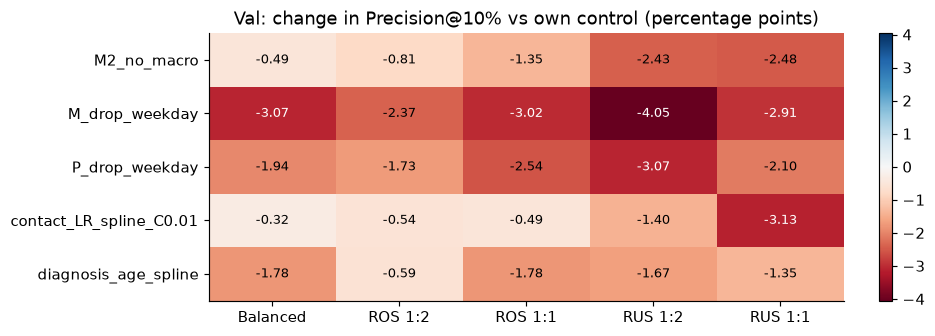

In [14]:
# Historical saved summary: percentage-point differences, not new fits.
delta=pd.DataFrame([[-0.4854368932038833, -0.8090614886731351, -1.3484358144552315, -2.4271844660194137, -2.481121898597624], [-3.0744336569579254, -2.3732470334412032, -3.0204962243797153, -4.045307443365692, -2.912621359223297], [-1.9417475728155305, -1.7259978425026967, -2.535059331175832, -3.0744336569579254, -2.103559870550159], [-0.32362459546925737, -0.5393743257820993, -0.48543689320388883, -1.402373247033445, -3.1283710895361416], [-1.7799352750809072, -0.5933117583603015, -1.7799352750809043, -1.6720604099244891, -1.3484358144552315]],
    index=['M2_no_macro', 'M_drop_weekday', 'P_drop_weekday', 'contact_LR_spline_C0.01', 'diagnosis_age_spline'],
    columns=['balanced', 'ros_1to2', 'ros_1to1', 'rus_1to2', 'rus_1to1'])
fig,ax=plt.subplots(figsize=(9,3.3))
bound=max(1.,float(np.abs(delta.to_numpy()).max()))
im=ax.imshow(delta,vmin=-bound,vmax=bound,cmap='RdBu',aspect='auto')
ax.set(xticks=np.arange(len(delta.columns)),xticklabels=['Balanced','ROS 1:2','ROS 1:1','RUS 1:2','RUS 1:1'],
       yticks=np.arange(len(delta)),yticklabels=delta.index,title='Val: change in Precision@10% vs own control (percentage points)')
for i in range(len(delta)):
    for j in range(len(delta.columns)):ax.text(j,i,f'{delta.iloc[i,j]:+.2f}',ha='center',va='center',fontsize=9,color='white' if abs(delta.iloc[i,j])>bound*.7 else 'black')
fig.colorbar(im,ax=ax,fraction=.04);finish(fig,'07_imbalance_paired')

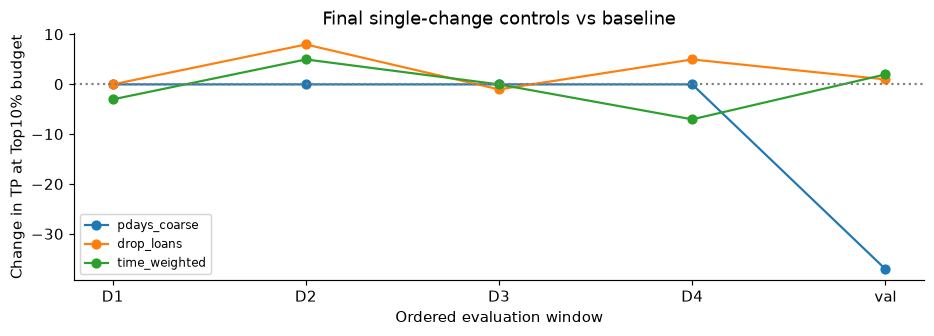

In [15]:
# Historical saved TP counts at a fixed Top10% budget.
variants=['baseline', 'pdays_coarse', 'drop_loans', 'time_weighted']
folds=['D1', 'D2', 'D3', 'D4', 'val']
pivot=pd.DataFrame([[29, 29, 29, 26], [19, 27, 19, 24], [17, 16, 17, 17], [63, 68, 63, 56], [172, 173, 135, 174]],index=folds,columns=['baseline', 'drop_loans', 'pdays_coarse', 'time_weighted'])
fig,ax=plt.subplots(figsize=(9,3.3))
for variant in variants[1:]:ax.plot(folds,pivot[variant]-pivot['baseline'],marker='o',label=variant)
ax.axhline(0,color='grey',ls=':');ax.set(ylabel='Change in TP at Top10% budget',xlabel='Ordered evaluation window',title='Final single-change controls vs baseline')
ax.legend(fontsize=8);finish(fig,'08_final_refinement')

### Optional original atlas / 原可选探索图集

保留原可选图集代码；图集属于描述与开发过程，不是补充模型的test性能表。



In [16]:
def display_groups(field):
    if field=='age':
        return [pd.cut(d[field],np.arange(15,105,5),right=False).astype(str) for d in [train,val]]
    if field in ['campaign','previous']:
        return [d[field].map(lambda x:str(x) if x<4 else '4+').astype(str) for d in [train,val]]
    if field=='pdays':
        return [pd.cut(d[field],[-np.inf,0,7,30,998,np.inf],
                       labels=['0','1–7','8–30','31–998','999']).astype(str) for d in [train,val]]
    if pd.api.types.is_numeric_dtype(train[field]):
        inside=np.unique(train[field].quantile([.25,.5,.75]).to_numpy())
        bins=np.r_[-np.inf,inside,np.inf]
        return [pd.cut(d[field],bins).astype(str) for d in [train,val]]
    return [d[field].astype(str) for d in [train,val]]

if SHOW_ALL_20_FIELDS:
    for field in train.columns.drop('y'):
        series=display_groups(field);fig,axes=plt.subplots(1,2,figsize=(10,4))
        counts=[]
        for split,d,g in zip(['train','val'],[train,val],series):
            tab=pd.DataFrame({'group':g,'yes':d.y.eq('yes').astype(int)}).groupby('group',sort=True).yes.agg(['size','mean'])
            axes[0].plot(tab.index,tab['mean']*100,marker='o',label=split,color=COLORS[split])
            axes[0].axhline(d.y.eq('yes').mean()*100,color=COLORS[split],ls=':',alpha=.6)
            if split=='val':axes[1].bar(tab.index,tab['size'],color=COLORS[split])
        axes[0].set(title=field,xlabel='Group',ylabel='Yes rate (%)');axes[0].legend()
        axes[1].set(title='Validation group size',ylabel='N')
        for ax in axes:ax.tick_params(axis='x',rotation=70)
        finish(fig,'optional_'+field)
else:
    print('Optional 20-field plots are off; set SHOW_ALL_20_FIELDS=True to regenerate from CSV.')


Optional 20-field plots are off; set SHOW_ALL_20_FIELDS=True to regenerate from CSV.


## 12. Final metric leaderboards / 各指标前5模型与冻结阶段

本节汇总此前已保存的 **同一份 test** 结果：行 `[35009, 41188)`，6,179 人、2,376 个 yes，正类率 38.4528%。这里的“前5”是**每项指标分别排序的描述性结果**，不据此选出新的最终模型，也不新增训练、预测或阈值搜索。原有 train/val 开发结果不混入本榜。

**冻结阶段如何看：**

| 表内标记 | 具体含义 | 证据边界 |
|---|---|---|
| 冻结前：首次冻结方案 | A、B、A_scaled，见第6节；A_scaled 原由 val 选定 | 首次冻结方案的 test 评价 |
| 冻结前开发；冻结后补测 | B_default3、B_macro_all、B_month、B_pdays 已出现在原开发比较，但不属于第6节首次测试的三个模型 | 后来的 test 补测，不能补称独立确认 |
| 冻结后：探索/补充评估 | 第7节起提出、调整或补充评价的方案，包括类权重、重采样、校准、窗口、时间权重和卡尔曼等 | `POSTHOC_SUPPLEMENTARY_TEST_NOT_INDEPENDENT_CONFIRMATION` |

“冻结后”不表示用 test 拟合；这些实验仍按各节记录在 train/val 拟合、调参或冻结规则。区别在于开发时已经知晓此前的 test 结果。

**覆盖与去重：** 407 条分节引用涉及275个预测标识；根据已保存完整预测文件的相同内容合并重复引用，得到 **226 个结果**。其中 **6 个常数参照**单列，主榜包含 **220 个模型/概率配置**。同一模型在多个章节反复出现只占一项；不同参数、随机种子或校准映射是不同配置。仅指标碰巧相同不合并。完整名称及别名在本节末折叠表中。

**排名口径：** ROC-AUC、AP 越大越好；Brier、Log loss、ECE10 越小越好。这5项不依赖分类阈值，仅展示一次。Accuracy、Precision、Recall、F1、Specificity、Balanced Accuracy、Lift 以及 TP/TN/FP/FN 分别按固定 Top10%、固定0.5、Top5%和Top20%排名。预算规则使用预设联系人数及原来的并列处理；不会按 test 标签重新取阈值。各支线不统一的 val F1/Recall 等已保存阈值仍留在原章节，不混进这些统一口径榜。

每表显示5个配置；按完整精度读入、保留12位小数判断并列，显示6位小数。并列用固定名称顺序决定展示次序，**不代表优劣**；第5条截断并列时可展开全部同分配置。未定义的 Precision/Lift 不参加相应排名。N、Yes、Yes rate、Threshold、Mean p、Contacts 是样本/操作描述，没有统一“越大越好”方向，不单独排名。TP/TN 越大、FP/FN 越小的榜只是分类结果的拆解，不是四个独立的选模目标。

下面的代码内嵌完整排名输入和计算逻辑；不依赖本机审计目录或额外 CSV。可从本节第一段代码依次重跑，仅重新排列表格。原主 Notebook 其他部分的执行行为保持原样。


In [ ]:
# Saved-result snapshot: no raw-data reads, fitting, prediction, or threshold search.
# This cell is self-contained and uses only the dependencies already used by this notebook.
from io import StringIO
from html import escape
import numpy as np
import pandas as pd
from IPython.display import HTML, display

TOP5_MODEL_CSV = r"""
model_id,model,phase,evidence,reference,aliases,alias_count,display_order
original__B_default3,B_default3,冻结前开发；冻结后补测,事后补测，非独立确认,False,closeout_test / original__B_default3,1,0
original__B_macro_all,B_macro_all,冻结前开发；冻结后补测,事后补测，非独立确认,False,closeout_test / original__B_macro_all,1,1
original__B_month,B_month,冻结前开发；冻结后补测,事后补测，非独立确认,False,closeout_test / original__B_month,1,2
original__B_pdays,B_pdays,冻结前开发；冻结后补测,事后补测，非独立确认,False,closeout_test / original__B_pdays,1,3
reference__train_prior,train_prior_dummy（常数）,冻结前：常数参照,第6节原始参照,True,closeout_test / reference__train_prior；diagnosis / train_prior_dummy；macro / train_prior_dummy；personal_macro / train_prior,4,4
original__A,A,冻结前：首次冻结方案,第6节首次test评估,False,closeout_test / original__A,1,5
original__A_scaled,A_scaled,冻结前：首次冻结方案,第6节首次test评估,False,closeout_test / diagnostic_reconstructed__baseline；closeout_test / original__A_scaled；diagnosis / baseline,3,6
original__B,B,冻结前：首次冻结方案,第6节首次test评估,False,closeout_test / original__B,1,7
boosting_error_audit__contact_HGB_d2_l21,HGB / contact_HGB_d2_l21,冻结后：探索/补充评估,事后探索，非独立确认,False,boosting / contact_HGB_d2_l21；closeout_test / boosting_error_audit__contact_HGB_d2_l21,2,8
boosting_error_audit__contact_HGB_d2_l210,HGB / contact_HGB_d2_l210,冻结后：探索/补充评估,事后探索，非独立确认,False,boosting / contact_HGB_d2_l210；closeout_test / boosting_error_audit__contact_HGB_d2_l210,2,9
boosting_error_audit__contact_HGB_d3_l21,HGB / contact_HGB_d3_l21,冻结后：探索/补充评估,事后探索，非独立确认,False,boosting / contact_HGB_d3_l21；closeout_test / boosting_error_audit__contact_HGB_d3_l21,2,10
boosting_error_audit__contact_HGB_d3_l210,HGB / contact_HGB_d3_l210,冻结后：探索/补充评估,事后探索，非独立确认,False,boosting / contact_HGB_d3_l210；closeout_test / boosting_error_audit__contact_HGB_d3_l210,2,11
boosting_error_audit__personal_HGB_d2_l21,HGB / personal_HGB_d2_l21,冻结后：探索/补充评估,事后探索，非独立确认,False,boosting / personal_HGB_d2_l21；closeout_test / boosting_error_audit__personal_HGB_d2_l21,2,12
boosting_error_audit__personal_HGB_d2_l210,HGB / personal_HGB_d2_l210,冻结后：探索/补充评估,事后探索，非独立确认,False,boosting / personal_HGB_d2_l210；closeout_test / boosting_error_audit__personal_HGB_d2_l210,2,13
boosting_error_audit__personal_HGB_d3_l21,HGB / personal_HGB_d3_l21,冻结后：探索/补充评估,事后探索，非独立确认,False,boosting / personal_HGB_d3_l21；closeout_test / boosting_error_audit__personal_HGB_d3_l21,2,14
boosting_error_audit__personal_HGB_d3_l210,HGB / personal_HGB_d3_l210,冻结后：探索/补充评估,事后探索，非独立确认,False,boosting / personal_HGB_d3_l210；closeout_test / boosting_error_audit__personal_HGB_d3_l210,2,15
test__M2_no_macro__balanced__0,不平衡处理 / M2_no_macro | balanced | seed=0,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M2_no_macro | balanced | seed=0,1,16
test__M2_no_macro__ros_1to1__17,不平衡处理 / M2_no_macro | ros_1to1 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M2_no_macro | ros_1to1 | seed=17,1,17
test__M2_no_macro__ros_1to1__2026,不平衡处理 / M2_no_macro | ros_1to1 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M2_no_macro | ros_1to1 | seed=2026,1,18
test__M2_no_macro__ros_1to1__42,不平衡处理 / M2_no_macro | ros_1to1 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M2_no_macro | ros_1to1 | seed=42,1,19
test__M2_no_macro__ros_1to2__17,不平衡处理 / M2_no_macro | ros_1to2 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M2_no_macro | ros_1to2 | seed=17,1,20
test__M2_no_macro__ros_1to2__2026,不平衡处理 / M2_no_macro | ros_1to2 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M2_no_macro | ros_1to2 | seed=2026,1,21
test__M2_no_macro__ros_1to2__42,不平衡处理 / M2_no_macro | ros_1to2 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M2_no_macro | ros_1to2 | seed=42,1,22
test__M2_no_macro__rus_1to1__17,不平衡处理 / M2_no_macro | rus_1to1 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M2_no_macro | rus_1to1 | seed=17,1,23
test__M2_no_macro__rus_1to1__2026,不平衡处理 / M2_no_macro | rus_1to1 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M2_no_macro | rus_1to1 | seed=2026,1,24
test__M2_no_macro__rus_1to1__42,不平衡处理 / M2_no_macro | rus_1to1 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M2_no_macro | rus_1to1 | seed=42,1,25
test__M2_no_macro__rus_1to2__17,不平衡处理 / M2_no_macro | rus_1to2 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M2_no_macro | rus_1to2 | seed=17,1,26
test__M2_no_macro__rus_1to2__2026,不平衡处理 / M2_no_macro | rus_1to2 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M2_no_macro | rus_1to2 | seed=2026,1,27
test__M2_no_macro__rus_1to2__42,不平衡处理 / M2_no_macro | rus_1to2 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M2_no_macro | rus_1to2 | seed=42,1,28
test__M_drop_weekday__balanced__0,不平衡处理 / M_drop_weekday | balanced | seed=0,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M_drop_weekday | balanced | seed=0,1,29
test__M_drop_weekday__ros_1to1__17,不平衡处理 / M_drop_weekday | ros_1to1 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M_drop_weekday | ros_1to1 | seed=17,1,30
test__M_drop_weekday__ros_1to1__2026,不平衡处理 / M_drop_weekday | ros_1to1 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M_drop_weekday | ros_1to1 | seed=2026,1,31
test__M_drop_weekday__ros_1to1__42,不平衡处理 / M_drop_weekday | ros_1to1 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M_drop_weekday | ros_1to1 | seed=42,1,32
test__M_drop_weekday__ros_1to2__17,不平衡处理 / M_drop_weekday | ros_1to2 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M_drop_weekday | ros_1to2 | seed=17,1,33
test__M_drop_weekday__ros_1to2__2026,不平衡处理 / M_drop_weekday | ros_1to2 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M_drop_weekday | ros_1to2 | seed=2026,1,34
test__M_drop_weekday__ros_1to2__42,不平衡处理 / M_drop_weekday | ros_1to2 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M_drop_weekday | ros_1to2 | seed=42,1,35
test__M_drop_weekday__rus_1to1__17,不平衡处理 / M_drop_weekday | rus_1to1 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M_drop_weekday | rus_1to1 | seed=17,1,36
test__M_drop_weekday__rus_1to1__2026,不平衡处理 / M_drop_weekday | rus_1to1 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M_drop_weekday | rus_1to1 | seed=2026,1,37
test__M_drop_weekday__rus_1to1__42,不平衡处理 / M_drop_weekday | rus_1to1 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M_drop_weekday | rus_1to1 | seed=42,1,38
test__M_drop_weekday__rus_1to2__17,不平衡处理 / M_drop_weekday | rus_1to2 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M_drop_weekday | rus_1to2 | seed=17,1,39
test__M_drop_weekday__rus_1to2__2026,不平衡处理 / M_drop_weekday | rus_1to2 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M_drop_weekday | rus_1to2 | seed=2026,1,40
test__M_drop_weekday__rus_1to2__42,不平衡处理 / M_drop_weekday | rus_1to2 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / M_drop_weekday | rus_1to2 | seed=42,1,41
test__P_drop_weekday__balanced__0,不平衡处理 / P_drop_weekday | balanced | seed=0,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / P_drop_weekday | balanced | seed=0,1,42
test__P_drop_weekday__ros_1to1__17,不平衡处理 / P_drop_weekday | ros_1to1 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / P_drop_weekday | ros_1to1 | seed=17,1,43
test__P_drop_weekday__ros_1to1__2026,不平衡处理 / P_drop_weekday | ros_1to1 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / P_drop_weekday | ros_1to1 | seed=2026,1,44
test__P_drop_weekday__ros_1to1__42,不平衡处理 / P_drop_weekday | ros_1to1 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / P_drop_weekday | ros_1to1 | seed=42,1,45
test__P_drop_weekday__ros_1to2__17,不平衡处理 / P_drop_weekday | ros_1to2 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / P_drop_weekday | ros_1to2 | seed=17,1,46
test__P_drop_weekday__ros_1to2__2026,不平衡处理 / P_drop_weekday | ros_1to2 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / P_drop_weekday | ros_1to2 | seed=2026,1,47
test__P_drop_weekday__ros_1to2__42,不平衡处理 / P_drop_weekday | ros_1to2 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / P_drop_weekday | ros_1to2 | seed=42,1,48
test__P_drop_weekday__rus_1to1__17,不平衡处理 / P_drop_weekday | rus_1to1 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / P_drop_weekday | rus_1to1 | seed=17,1,49
test__P_drop_weekday__rus_1to1__2026,不平衡处理 / P_drop_weekday | rus_1to1 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / P_drop_weekday | rus_1to1 | seed=2026,1,50
test__P_drop_weekday__rus_1to1__42,不平衡处理 / P_drop_weekday | rus_1to1 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / P_drop_weekday | rus_1to1 | seed=42,1,51
test__P_drop_weekday__rus_1to2__17,不平衡处理 / P_drop_weekday | rus_1to2 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / P_drop_weekday | rus_1to2 | seed=17,1,52
test__P_drop_weekday__rus_1to2__2026,不平衡处理 / P_drop_weekday | rus_1to2 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / P_drop_weekday | rus_1to2 | seed=2026,1,53
test__P_drop_weekday__rus_1to2__42,不平衡处理 / P_drop_weekday | rus_1to2 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / P_drop_weekday | rus_1to2 | seed=42,1,54
test__contact_LR_spline_C0.01__balanced__0,不平衡处理 / contact_LR_spline_C0.01 | balanced | seed=0,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_W | E | raw；calibration / LR_W | S | raw；calibration / LR_W | W | raw；history_diagnostic / LR_W；imbalance / contact_LR_spline_C0.01 | balanced | seed=0,5,55
test__contact_LR_spline_C0.01__balanced_rf__17,不平衡处理 / contact_LR_spline_C0.01 | balanced_rf | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | balanced_rf | seed=17,1,56
test__contact_LR_spline_C0.01__balanced_rf__2026,不平衡处理 / contact_LR_spline_C0.01 | balanced_rf | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | balanced_rf | seed=2026,1,57
test__contact_LR_spline_C0.01__balanced_rf__42,不平衡处理 / contact_LR_spline_C0.01 | balanced_rf | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | balanced_rf | seed=42,1,58
test__contact_LR_spline_C0.01__ordinary_rf__17,不平衡处理 / contact_LR_spline_C0.01 | ordinary_rf | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | ordinary_rf | seed=17,1,59
test__contact_LR_spline_C0.01__ordinary_rf__2026,不平衡处理 / contact_LR_spline_C0.01 | ordinary_rf | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | ordinary_rf | seed=2026,1,60
test__contact_LR_spline_C0.01__ordinary_rf__42,不平衡处理 / contact_LR_spline_C0.01 | ordinary_rf | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / RF | E | raw；calibration / RF | S | raw；calibration / RF | W | raw；history_diagnostic / RF；imbalance / contact_LR_spline_C0.01 | ordinary_rf | seed=42；window / RF | full_history,6,61
test__contact_LR_spline_C0.01__ros_1to1__17,不平衡处理 / contact_LR_spline_C0.01 | ros_1to1 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | ros_1to1 | seed=17,1,62
test__contact_LR_spline_C0.01__ros_1to1__2026,不平衡处理 / contact_LR_spline_C0.01 | ros_1to1 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | ros_1to1 | seed=2026,1,63
test__contact_LR_spline_C0.01__ros_1to1__42,不平衡处理 / contact_LR_spline_C0.01 | ros_1to1 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | ros_1to1 | seed=42,1,64
test__contact_LR_spline_C0.01__ros_1to2__17,不平衡处理 / contact_LR_spline_C0.01 | ros_1to2 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | ros_1to2 | seed=17,1,65
test__contact_LR_spline_C0.01__ros_1to2__2026,不平衡处理 / contact_LR_spline_C0.01 | ros_1to2 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | ros_1to2 | seed=2026,1,66
test__contact_LR_spline_C0.01__ros_1to2__42,不平衡处理 / contact_LR_spline_C0.01 | ros_1to2 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_O2 | E | raw；calibration / LR_O2 | S | raw；calibration / LR_O2 | W | raw；history_diagnostic / LR_O2；imbalance / contact_LR_spline_C0.01 | ros_1to2 | seed=42,5,67
test__contact_LR_spline_C0.01__rus_1to1__17,不平衡处理 / contact_LR_spline_C0.01 | rus_1to1 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | rus_1to1 | seed=17,1,68
test__contact_LR_spline_C0.01__rus_1to1__2026,不平衡处理 / contact_LR_spline_C0.01 | rus_1to1 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | rus_1to1 | seed=2026,1,69
test__contact_LR_spline_C0.01__rus_1to1__42,不平衡处理 / contact_LR_spline_C0.01 | rus_1to1 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | rus_1to1 | seed=42,1,70
test__contact_LR_spline_C0.01__rus_1to2__17,不平衡处理 / contact_LR_spline_C0.01 | rus_1to2 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | rus_1to2 | seed=17,1,71
test__contact_LR_spline_C0.01__rus_1to2__2026,不平衡处理 / contact_LR_spline_C0.01 | rus_1to2 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | rus_1to2 | seed=2026,1,72
test__contact_LR_spline_C0.01__rus_1to2__42,不平衡处理 / contact_LR_spline_C0.01 | rus_1to2 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | rus_1to2 | seed=42,1,73
test__contact_LR_spline_C0.01__weighted_rf__17,不平衡处理 / contact_LR_spline_C0.01 | weighted_rf | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | weighted_rf | seed=17,1,74
test__contact_LR_spline_C0.01__weighted_rf__2026,不平衡处理 / contact_LR_spline_C0.01 | weighted_rf | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | weighted_rf | seed=2026,1,75
test__contact_LR_spline_C0.01__weighted_rf__42,不平衡处理 / contact_LR_spline_C0.01 | weighted_rf | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / contact_LR_spline_C0.01 | weighted_rf | seed=42,1,76
test__diagnosis_age_spline__balanced__0,不平衡处理 / diagnosis_age_spline | balanced | seed=0,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / diagnosis_age_spline | balanced | seed=0,1,77
test__diagnosis_age_spline__ros_1to1__17,不平衡处理 / diagnosis_age_spline | ros_1to1 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / diagnosis_age_spline | ros_1to1 | seed=17,1,78
test__diagnosis_age_spline__ros_1to1__2026,不平衡处理 / diagnosis_age_spline | ros_1to1 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / diagnosis_age_spline | ros_1to1 | seed=2026,1,79
test__diagnosis_age_spline__ros_1to1__42,不平衡处理 / diagnosis_age_spline | ros_1to1 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / diagnosis_age_spline | ros_1to1 | seed=42,1,80
test__diagnosis_age_spline__ros_1to2__17,不平衡处理 / diagnosis_age_spline | ros_1to2 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / diagnosis_age_spline | ros_1to2 | seed=17,1,81
test__diagnosis_age_spline__ros_1to2__2026,不平衡处理 / diagnosis_age_spline | ros_1to2 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / diagnosis_age_spline | ros_1to2 | seed=2026,1,82
test__diagnosis_age_spline__ros_1to2__42,不平衡处理 / diagnosis_age_spline | ros_1to2 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / diagnosis_age_spline | ros_1to2 | seed=42,1,83
test__diagnosis_age_spline__rus_1to1__17,不平衡处理 / diagnosis_age_spline | rus_1to1 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / diagnosis_age_spline | rus_1to1 | seed=17,1,84
test__diagnosis_age_spline__rus_1to1__2026,不平衡处理 / diagnosis_age_spline | rus_1to1 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / diagnosis_age_spline | rus_1to1 | seed=2026,1,85
test__diagnosis_age_spline__rus_1to1__42,不平衡处理 / diagnosis_age_spline | rus_1to1 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / diagnosis_age_spline | rus_1to1 | seed=42,1,86
test__diagnosis_age_spline__rus_1to2__17,不平衡处理 / diagnosis_age_spline | rus_1to2 | seed=17,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / diagnosis_age_spline | rus_1to2 | seed=17,1,87
test__diagnosis_age_spline__rus_1to2__2026,不平衡处理 / diagnosis_age_spline | rus_1to2 | seed=2026,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / diagnosis_age_spline | rus_1to2 | seed=2026,1,88
test__diagnosis_age_spline__rus_1to2__42,不平衡处理 / diagnosis_age_spline | rus_1to2 | seed=42,冻结后：探索/补充评估,事后探索，非独立确认,False,imbalance / diagnosis_age_spline | rus_1to2 | seed=42,1,89
diagnostic_reconstructed__age_spline_strict,严格求解 / age_spline_strict,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / diagnostic_reconstructed__age_spline_strict；diagnosis_followup / age_spline_strict；history_diagnostic / diagnosis_age_spline；imbalance / diagnosis_age_spline | none | seed=0,4,90
personal_macro_v2__M_drop_age,个人/联系/宏观设计 / M_drop_age,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__M_drop_age；personal_macro / M_drop_age,2,91
personal_macro_v2__M_drop_campaign,个人/联系/宏观设计 / M_drop_campaign,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__M_drop_campaign；personal_macro / M_drop_campaign,2,92
personal_macro_v2__M_drop_contact,个人/联系/宏观设计 / M_drop_contact,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__M_drop_contact；personal_macro / M_drop_contact,2,93
personal_macro_v2__M_drop_default,个人/联系/宏观设计 / M_drop_default,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__M_drop_default；personal_macro / M_drop_default,2,94
personal_macro_v2__M_drop_education,个人/联系/宏观设计 / M_drop_education,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__M_drop_education；personal_macro / M_drop_education,2,95
personal_macro_v2__M_drop_history,个人/联系/宏观设计 / M_drop_history,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__M_drop_history；personal_macro / M_drop_history,2,96
personal_macro_v2__M_drop_job,个人/联系/宏观设计 / M_drop_job,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__M_drop_job；personal_macro / M_drop_job,2,97
personal_macro_v2__M_drop_loans,个人/联系/宏观设计 / M_drop_loans,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__M_drop_loans；personal_macro / M_drop_loans,2,98
personal_macro_v2__M_drop_marital,个人/联系/宏观设计 / M_drop_marital,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__M_drop_marital；personal_macro / M_drop_marital,2,99
personal_macro_v2__M_drop_month,个人/联系/宏观设计 / M_drop_month,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__M_drop_month；personal_macro / M_drop_month,2,100
personal_macro_v2__M_drop_weekday,个人/联系/宏观设计 / M_drop_weekday,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__M_drop_weekday；history_diagnostic / M_drop_weekday；imbalance / M_drop_weekday | none | seed=0；personal_macro / M_drop_weekday；personal_macro_test / M_drop_weekday,5,101
personal_macro_v2__M_penalty1,个人/联系/宏观设计 / M_penalty1,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__M_penalty1；personal_macro / M_penalty1；personal_macro_test / M_penalty1,3,102
personal_macro_v2__M_penalty10,个人/联系/宏观设计 / M_penalty10,冻结后：探索/补充评估,事后探索，非独立确认,False,binning / M_penalty10__current；closeout_test / personal_macro_v2__M_penalty10；closeout_test / weight_interaction__M10_w1_i0；personal_macro / M_penalty10；personal_macro_test / M_penalty10；weights / M10_w1_i0,6,103
personal_macro_v2__M_penalty100,个人/联系/宏观设计 / M_penalty100,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__M_penalty100；personal_macro / M_penalty100；personal_macro_test / M_penalty100,3,104
personal_macro_v2__P0_linear,个人/联系/宏观设计 / P0_linear,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__P0_linear；personal_macro / P0_linear；personal_macro_test / P0_linear,3,105
personal_macro_v2__P1_age_spline,个人/联系/宏观设计 / P1_age_spline,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__P1_age_spline；personal_macro / P1_age_spline；personal_macro_test / P1_age_spline,3,106
personal_macro_v2__P2_previous,个人/联系/宏观设计 / P2_previous,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__P2_previous；personal_macro / P2_previous；personal_macro_test / P2_previous,3,107
personal_macro_v2__P3_pdays_flag,个人/联系/宏观设计 / P3_pdays_flag,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__P3_pdays_flag；personal_macro / P3_pdays_flag；personal_macro_test / P3_pdays_flag,3,108
personal_macro_v2__P_drop_age,个人/联系/宏观设计 / P_drop_age,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__P_drop_age；personal_macro / P_drop_age,2,109
personal_macro_v2__P_drop_campaign,个人/联系/宏观设计 / P_drop_campaign,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__P_drop_campaign；personal_macro / P_drop_campaign,2,110
personal_macro_v2__P_drop_contact,个人/联系/宏观设计 / P_drop_contact,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__P_drop_contact；personal_macro / P_drop_contact,2,111
personal_macro_v2__P_drop_default,个人/联系/宏观设计 / P_drop_default,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__P_drop_default；personal_macro / P_drop_default,2,112
personal_macro_v2__P_drop_education,个人/联系/宏观设计 / P_drop_education,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__P_drop_education；personal_macro / P_drop_education,2,113
personal_macro_v2__P_drop_history,个人/联系/宏观设计 / P_drop_history,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__P_drop_history；personal_macro / P_drop_history,2,114
personal_macro_v2__P_drop_job,个人/联系/宏观设计 / P_drop_job,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__P_drop_job；personal_macro / P_drop_job,2,115
personal_macro_v2__P_drop_loans,个人/联系/宏观设计 / P_drop_loans,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__P_drop_loans；personal_macro / P_drop_loans,2,116
personal_macro_v2__P_drop_marital,个人/联系/宏观设计 / P_drop_marital,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__P_drop_marital；personal_macro / P_drop_marital,2,117
personal_macro_v2__P_drop_month,个人/联系/宏观设计 / P_drop_month,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__P_drop_month；personal_macro / P_drop_month,2,118
personal_macro_v2__P_drop_weekday,个人/联系/宏观设计 / P_drop_weekday,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / personal_macro_v2__P_drop_weekday；history_diagnostic / P_drop_weekday；imbalance / P_drop_weekday | none | seed=0；personal_macro / P_drop_weekday；personal_macro_test / P_drop_weekday,5,119
personal_macro_v2__P_full,个人/联系/宏观设计 / P_full,冻结后：探索/补充评估,事后探索，非独立确认,False,binning / P_full__current；closeout_test / personal_macro_v2__P_full；closeout_test / weight_interaction__P_w1_i0；personal_macro / P_full；personal_macro_test / P_full；weights / P_w1_i0,6,120
information_scope__personal_contact_history,信息范围 / personal_contact_history,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / information_scope__personal_contact_history；closeout_test / precision_constraints__contact_LR_spline_C1；precision / contact_LR_spline_C1；precision / personal_contact_history；scope / personal_contact_history,5,121
information_scope__personal_only,信息范围 / personal_only,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / information_scope__personal_only；closeout_test / precision_constraints__personal_LR_spline_C1；precision / personal_LR_spline_C1；precision / personal_only；scope / personal_only,5,122
new_binning__M_penalty10__both,分箱 / M_penalty10__both,冻结后：探索/补充评估,事后探索，非独立确认,False,binning / M_penalty10__both,1,123
new_binning__M_penalty10__campaign_only,分箱 / M_penalty10__campaign_only,冻结后：探索/补充评估,事后探索，非独立确认,False,binning / M_penalty10__campaign_only,1,124
new_binning__M_penalty10__pdays_only,分箱 / M_penalty10__pdays_only,冻结后：探索/补充评估,事后探索，非独立确认,False,binning / M_penalty10__pdays_only,1,125
new_binning__P_full__both,分箱 / P_full__both,冻结后：探索/补充评估,事后探索，非独立确认,False,binning / P_full__both,1,126
new_binning__P_full__campaign_only,分箱 / P_full__campaign_only,冻结后：探索/补充评估,事后探索，非独立确认,False,binning / P_full__campaign_only,1,127
new_binning__P_full__pdays_only,分箱 / P_full__pdays_only,冻结后：探索/补充评估,事后探索，非独立确认,False,binning / P_full__pdays_only,1,128
calibration__LR_N__E__intercept_only,前向概率校准 / LR_N | E | intercept_only,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_N | E | intercept_only,1,129
calibration__LR_N__E__prior_natural,前向概率校准 / LR_N | E | prior_natural,冻结后：探索/补充评估,事后探索，非独立确认,True,calibration / LR_N | E | prior_natural；calibration / LR_N | E | prior_weighted；calibration / LR_N | W | prior_natural；calibration / LR_O2 | E | prior_natural；calibration / LR_O2 | E | prior_weighted；calibration / LR_O2 | W | prior_natural；calibration / LR_W | E | prior_natural；calibration / LR_W | E | prior_weighted；calibration / LR_W | W | prior_natural；calibration / RF | E | prior_natural；calibration / RF | E | prior_weighted；calibration / RF | W | prior_natural,12,130
calibration__LR_N__E__sigmoid_positive_slope,前向概率校准 / LR_N | E | sigmoid_positive_slope,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_N | E | sigmoid_positive_slope,1,131
calibration__LR_N__S__intercept_only,前向概率校准 / LR_N | S | intercept_only,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_N | S | intercept_only,1,132
calibration__LR_N__S__prior_natural,前向概率校准 / LR_N | S | prior_natural,冻结后：探索/补充评估,事后探索，非独立确认,True,calibration / LR_N | S | prior_natural；calibration / LR_N | S | prior_weighted；calibration / LR_O2 | S | prior_natural；calibration / LR_O2 | S | prior_weighted；calibration / LR_W | S | prior_natural；calibration / LR_W | S | prior_weighted；calibration / RF | S | prior_natural；calibration / RF | S | prior_weighted,8,133
calibration__LR_N__S__sigmoid_positive_slope,前向概率校准 / LR_N | S | sigmoid_positive_slope,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_N | S | sigmoid_positive_slope,1,134
calibration__LR_N__W__intercept_only,前向概率校准 / LR_N | W | intercept_only,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_N | W | intercept_only,1,135
calibration__LR_N__W__prior_weighted,前向概率校准 / LR_N | W | prior_weighted,冻结后：探索/补充评估,事后探索，非独立确认,True,calibration / LR_N | W | prior_weighted；calibration / LR_O2 | W | prior_weighted；calibration / LR_W | W | prior_weighted；calibration / RF | W | prior_weighted,4,136
calibration__LR_N__W__sigmoid_positive_slope,前向概率校准 / LR_N | W | sigmoid_positive_slope,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_N | W | sigmoid_positive_slope,1,137
calibration__LR_O2__E__intercept_only,前向概率校准 / LR_O2 | E | intercept_only,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_O2 | E | intercept_only,1,138
calibration__LR_O2__E__sigmoid_positive_slope,前向概率校准 / LR_O2 | E | sigmoid_positive_slope,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_O2 | E | sigmoid_positive_slope,1,139
calibration__LR_O2__S__intercept_only,前向概率校准 / LR_O2 | S | intercept_only,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_O2 | S | intercept_only,1,140
calibration__LR_O2__S__sigmoid_positive_slope,前向概率校准 / LR_O2 | S | sigmoid_positive_slope,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_O2 | S | sigmoid_positive_slope,1,141
calibration__LR_O2__W__intercept_only,前向概率校准 / LR_O2 | W | intercept_only,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_O2 | W | intercept_only,1,142
calibration__LR_O2__W__sigmoid_positive_slope,前向概率校准 / LR_O2 | W | sigmoid_positive_slope,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_O2 | W | sigmoid_positive_slope,1,143
calibration__LR_W__E__intercept_only,前向概率校准 / LR_W | E | intercept_only,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_W | E | intercept_only,1,144
calibration__LR_W__E__sigmoid_positive_slope,前向概率校准 / LR_W | E | sigmoid_positive_slope,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_W | E | sigmoid_positive_slope,1,145
calibration__LR_W__S__intercept_only,前向概率校准 / LR_W | S | intercept_only,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_W | S | intercept_only,1,146
calibration__LR_W__S__sigmoid_positive_slope,前向概率校准 / LR_W | S | sigmoid_positive_slope,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_W | S | sigmoid_positive_slope,1,147
calibration__LR_W__W__intercept_only,前向概率校准 / LR_W | W | intercept_only,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_W | W | intercept_only,1,148
calibration__LR_W__W__sigmoid_positive_slope,前向概率校准 / LR_W | W | sigmoid_positive_slope,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_W | W | sigmoid_positive_slope,1,149
calibration__RF__E__intercept_only,前向概率校准 / RF | E | intercept_only,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / RF | E | intercept_only,1,150
calibration__RF__E__sigmoid_positive_slope,前向概率校准 / RF | E | sigmoid_positive_slope,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / RF | E | sigmoid_positive_slope,1,151
calibration__RF__S__intercept_only,前向概率校准 / RF | S | intercept_only,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / RF | S | intercept_only,1,152
calibration__RF__S__sigmoid_positive_slope,前向概率校准 / RF | S | sigmoid_positive_slope,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / RF | S | sigmoid_positive_slope,1,153
calibration__RF__W__intercept_only,前向概率校准 / RF | W | intercept_only,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / RF | W | intercept_only,1,154
calibration__RF__W__sigmoid_positive_slope,前向概率校准 / RF | W | sigmoid_positive_slope,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / RF | W | sigmoid_positive_slope,1,155
kalman__ewma,动态截距 / ewma,冻结后：探索/补充评估,事后探索，非独立确认,False,kalman / ewma,1,156
kalman__fixed_intercept,动态截距 / fixed_intercept,冻结后：探索/补充评估,事后探索，非独立确认,False,kalman / fixed_intercept,1,157
kalman__kalman,动态截距 / kalman,冻结后：探索/补充评估,事后探索，非独立确认,False,kalman / kalman,1,158
new_scale__poutcome_scale0.5,历史结果尺度 / poutcome_scale0.5,冻结后：探索/补充评估,事后探索，非独立确认,False,history_scale / poutcome_scale0.5,1,159
new_scale__poutcome_scale2.0,历史结果尺度 / poutcome_scale2.0,冻结后：探索/补充评估,事后探索，非独立确认,False,history_scale / poutcome_scale2.0,1,160
macro__M1_all_macro,宏观消融 / M1_all_macro,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / macro__M1_all_macro；macro / M1_all_macro；macro_test / M1_all_macro,3,161
macro__M2_no_macro,宏观消融 / M2_no_macro,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / macro__M2_no_macro；history_diagnostic / M2_no_macro；imbalance / M2_no_macro | none | seed=0；macro / M2_no_macro；macro_test / M2_no_macro,5,162
macro__M3_three_macro,宏观消融 / M3_three_macro,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / macro__M3_three_macro；macro / M3_three_macro；macro_test / M3_three_macro,3,163
temporal_calibration__M100__intercept_only,早期时间校准 / M100__intercept_only,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / temporal_calibration__M100__intercept_only；early_calibration / M100__intercept_only,2,164
temporal_calibration__M100__raw,早期时间校准 / M100__raw,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / temporal_calibration__M100__raw；early_calibration / M100__raw,2,165
temporal_calibration__M100__sigmoid_positive_slope,早期时间校准 / M100__sigmoid_positive_slope,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / temporal_calibration__M100__sigmoid_positive_slope；early_calibration / M100__sigmoid_positive_slope,2,166
temporal_calibration__M10__intercept_only,早期时间校准 / M10__intercept_only,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / temporal_calibration__M10__intercept_only；early_calibration / M10__intercept_only,2,167
temporal_calibration__M10__raw,早期时间校准 / M10__raw,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / temporal_calibration__M10__raw；early_calibration / M10__raw,2,168
temporal_calibration__M10__sigmoid_positive_slope,早期时间校准 / M10__sigmoid_positive_slope,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / temporal_calibration__M10__sigmoid_positive_slope；early_calibration / M10__sigmoid_positive_slope,2,169
temporal_calibration__P__intercept_only,早期时间校准 / P__intercept_only,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / temporal_calibration__P__intercept_only；early_calibration / P__intercept_only,2,170
temporal_calibration__P__raw,早期时间校准 / P__raw,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / temporal_calibration__P__raw；closeout_test / temporal_calibration__P__sigmoid_positive_slope；early_calibration / P__raw；early_calibration / P__sigmoid_positive_slope,4,171
new_refinement__drop_loans,最终小范围改进 / drop_loans,冻结后：探索/补充评估,事后探索，非独立确认,False,refinement / drop_loans,1,172
new_refinement__pdays_coarse,最终小范围改进 / pdays_coarse,冻结后：探索/补充评估,事后探索，非独立确认,False,refinement / pdays_coarse,1,173
new_refinement__time_weighted,最终小范围改进 / time_weighted,冻结后：探索/补充评估,事后探索，非独立确认,False,refinement / time_weighted,1,174
diagnostic_reconstructed__C_0.1,求解/表示诊断 / C_0.1,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / diagnostic_reconstructed__C_0.1；diagnosis / C_0.1,2,175
diagnostic_reconstructed__C_10,求解/表示诊断 / C_10,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / diagnostic_reconstructed__C_10；diagnosis / C_10,2,176
diagnostic_reconstructed__age_spline,求解/表示诊断 / age_spline,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / diagnostic_reconstructed__age_spline；diagnosis / age_spline,2,177
diagnostic_reconstructed__log_counts,求解/表示诊断 / log_counts,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / diagnostic_reconstructed__log_counts；diagnosis / log_counts,2,178
diagnostic_reconstructed__log_counts_age_spline,求解/表示诊断 / log_counts_age_spline,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / diagnostic_reconstructed__log_counts_age_spline；diagnosis / log_counts_age_spline,2,179
diagnostic_reconstructed__recent_12000,求解/表示诊断 / recent_12000,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / diagnostic_reconstructed__recent_12000；diagnosis / recent_12000,2,180
weight_interaction__M10_w1_i1,类权重/交互 / M10_w1_i1,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / weight_interaction__M10_w1_i1；weights / M10_w1_i1,2,181
weight_interaction__M10_w2_i0,类权重/交互 / M10_w2_i0,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / weight_interaction__M10_w2_i0；weights / M10_w2_i0,2,182
weight_interaction__M10_w2_i1,类权重/交互 / M10_w2_i1,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / weight_interaction__M10_w2_i1；weights / M10_w2_i1,2,183
weight_interaction__M10_w5_i0,类权重/交互 / M10_w5_i0,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / weight_interaction__M10_w5_i0；weights / M10_w5_i0,2,184
weight_interaction__M10_w5_i1,类权重/交互 / M10_w5_i1,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / weight_interaction__M10_w5_i1；weights / M10_w5_i1,2,185
weight_interaction__M10_wbalanced_i0,类权重/交互 / M10_wbalanced_i0,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / weight_interaction__M10_wbalanced_i0；weights / M10_wbalanced_i0,2,186
weight_interaction__M10_wbalanced_i1,类权重/交互 / M10_wbalanced_i1,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / weight_interaction__M10_wbalanced_i1；weights / M10_wbalanced_i1,2,187
weight_interaction__P_w1_i1,类权重/交互 / P_w1_i1,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / weight_interaction__P_w1_i1；weights / P_w1_i1,2,188
weight_interaction__P_w2_i0,类权重/交互 / P_w2_i0,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / weight_interaction__P_w2_i0；weights / P_w2_i0,2,189
weight_interaction__P_w2_i1,类权重/交互 / P_w2_i1,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / weight_interaction__P_w2_i1；weights / P_w2_i1,2,190
weight_interaction__P_w5_i0,类权重/交互 / P_w5_i0,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / weight_interaction__P_w5_i0；weights / P_w5_i0,2,191
weight_interaction__P_w5_i1,类权重/交互 / P_w5_i1,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / weight_interaction__P_w5_i1；weights / P_w5_i1,2,192
weight_interaction__P_wbalanced_i0,类权重/交互 / P_wbalanced_i0,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / weight_interaction__P_wbalanced_i0；weights / P_wbalanced_i0,2,193
weight_interaction__P_wbalanced_i1,类权重/交互 / P_wbalanced_i1,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / weight_interaction__P_wbalanced_i1；weights / P_wbalanced_i1,2,194
precision_constraints__contact_LR_linear_C0.01,联系模型/浅树 / contact_LR_linear_C0.01,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__contact_LR_linear_C0.01；precision / contact_LR_linear_C0.01,2,195
precision_constraints__contact_LR_linear_C0.1,联系模型/浅树 / contact_LR_linear_C0.1,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__contact_LR_linear_C0.1；precision / contact_LR_linear_C0.1,2,196
precision_constraints__contact_LR_linear_C1,联系模型/浅树 / contact_LR_linear_C1,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__contact_LR_linear_C1；precision / contact_LR_linear_C1,2,197
precision_constraints__contact_LR_linear_C10,联系模型/浅树 / contact_LR_linear_C10,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__contact_LR_linear_C10；precision / contact_LR_linear_C10,2,198
precision_constraints__contact_LR_spline_C0.01,联系模型/浅树 / contact_LR_spline_C0.01,冻结后：探索/补充评估,事后探索，非独立确认,False,calibration / LR_N | E | raw；calibration / LR_N | S | raw；calibration / LR_N | W | raw；closeout_test / precision_constraints__contact_LR_spline_C0.01；contact / contact_LR_spline_C0.01；history_diagnostic / LR_N；history_scale / poutcome_scale1.0；imbalance / contact_LR_spline_C0.01 | none | seed=0；kalman / raw；precision / contact_LR_spline_C0.01；refinement / baseline,11,199
precision_constraints__contact_LR_spline_C0.1,联系模型/浅树 / contact_LR_spline_C0.1,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__contact_LR_spline_C0.1；precision / contact_LR_spline_C0.1,2,200
precision_constraints__contact_LR_spline_C10,联系模型/浅树 / contact_LR_spline_C10,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__contact_LR_spline_C10；precision / contact_LR_spline_C10,2,201
precision_constraints__contact_TREE_d2_leaf100,联系模型/浅树 / contact_TREE_d2_leaf100,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__contact_TREE_d2_leaf100；precision / contact_TREE_d2_leaf100,2,202
precision_constraints__contact_TREE_d2_leaf300,联系模型/浅树 / contact_TREE_d2_leaf300,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__contact_TREE_d2_leaf300；precision / contact_TREE_d2_leaf300,2,203
precision_constraints__contact_TREE_d3_leaf100,联系模型/浅树 / contact_TREE_d3_leaf100,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__contact_TREE_d3_leaf100；precision / contact_TREE_d3_leaf100,2,204
precision_constraints__contact_TREE_d3_leaf300,联系模型/浅树 / contact_TREE_d3_leaf300,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__contact_TREE_d3_leaf300；precision / contact_TREE_d3_leaf300,2,205
precision_constraints__contact_TREE_d4_leaf100,联系模型/浅树 / contact_TREE_d4_leaf100,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__contact_TREE_d4_leaf100；precision / contact_TREE_d4_leaf100,2,206
precision_constraints__contact_TREE_d4_leaf300,联系模型/浅树 / contact_TREE_d4_leaf300,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__contact_TREE_d4_leaf300；precision / contact_TREE_d4_leaf300,2,207
precision_constraints__personal_LR_linear_C0.01,联系模型/浅树 / personal_LR_linear_C0.01,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__personal_LR_linear_C0.01；precision / personal_LR_linear_C0.01,2,208
precision_constraints__personal_LR_linear_C0.1,联系模型/浅树 / personal_LR_linear_C0.1,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__personal_LR_linear_C0.1；precision / personal_LR_linear_C0.1,2,209
precision_constraints__personal_LR_linear_C1,联系模型/浅树 / personal_LR_linear_C1,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__personal_LR_linear_C1；precision / personal_LR_linear_C1,2,210
precision_constraints__personal_LR_linear_C10,联系模型/浅树 / personal_LR_linear_C10,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__personal_LR_linear_C10；precision / personal_LR_linear_C10,2,211
precision_constraints__personal_LR_spline_C0.01,联系模型/浅树 / personal_LR_spline_C0.01,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__personal_LR_spline_C0.01；precision / personal_LR_spline_C0.01,2,212
precision_constraints__personal_LR_spline_C0.1,联系模型/浅树 / personal_LR_spline_C0.1,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__personal_LR_spline_C0.1；precision / personal_LR_spline_C0.1,2,213
precision_constraints__personal_LR_spline_C10,联系模型/浅树 / personal_LR_spline_C10,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__personal_LR_spline_C10；precision / personal_LR_spline_C10,2,214
precision_constraints__personal_TREE_d2_leaf100,联系模型/浅树 / personal_TREE_d2_leaf100,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__personal_TREE_d2_leaf100；precision / personal_TREE_d2_leaf100,2,215
precision_constraints__personal_TREE_d2_leaf300,联系模型/浅树 / personal_TREE_d2_leaf300,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__personal_TREE_d2_leaf300；precision / personal_TREE_d2_leaf300,2,216
precision_constraints__personal_TREE_d3_leaf100,联系模型/浅树 / personal_TREE_d3_leaf100,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__personal_TREE_d3_leaf100；precision / personal_TREE_d3_leaf100,2,217
precision_constraints__personal_TREE_d3_leaf300,联系模型/浅树 / personal_TREE_d3_leaf300,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__personal_TREE_d3_leaf300；precision / personal_TREE_d3_leaf300,2,218
precision_constraints__personal_TREE_d4_leaf100,联系模型/浅树 / personal_TREE_d4_leaf100,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__personal_TREE_d4_leaf100；precision / personal_TREE_d4_leaf100,2,219
precision_constraints__personal_TREE_d4_leaf300,联系模型/浅树 / personal_TREE_d4_leaf300,冻结后：探索/补充评估,事后探索，非独立确认,False,closeout_test / precision_constraints__personal_TREE_d4_leaf300；precision / personal_TREE_d4_leaf300,2,220
reference__all_no,补充评估 / reference__all_no,冻结后：探索/补充评估,事后探索，非独立确认,True,closeout_test / reference__all_no,1,221
reference__all_yes,补充评估 / reference__all_yes,冻结后：探索/补充评估,事后探索，非独立确认,True,closeout_test / reference__all_yes,1,222
new_window__HGB_val_full_history,近期窗口 / HGB | full_history,冻结后：探索/补充评估,事后探索，非独立确认,False,window / HGB | full_history,1,223
new_window__HGB_val_recent_12000,近期窗口 / HGB | recent_12000,冻结后：探索/补充评估,事后探索，非独立确认,False,window / HGB | recent_12000,1,224
new_window__RF_val_recent_12000,近期窗口 / RF | recent_12000,冻结后：探索/补充评估,事后探索，非独立确认,False,window / RF | recent_12000,1,225
"""
TOP5_METRIC_CSV = r"""
model_id,rule,n,yes,positive_rate,threshold,mean_probability,selected_n,precision_defined,roc_auc,average_precision,brier,log_loss,ece,accuracy,precision,recall,f1,specificity,balanced_accuracy,lift,tp,tn,fp,fn
original__A,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1853726318272598,362,True,0.5632119357303422,0.43978309375473046,0.2843369946999118,0.8365607335363504,0.2213553489534754,0.612558666450882,0.47513812154696133,0.0723905723905724,0.1256391526661797,0.9500394425453589,0.5112150074679657,1.2356390795617316,172,3613,190,2204
original__A,top5,6179,2376,0.38452824081566594,,0.1853726318272598,309,True,0.5632119357303422,0.43978309375473046,0.2843369946999118,0.8365607335363504,0.2213553489534754,0.6156335976695259,0.5016181229773463,0.06523569023569023,0.1154562383612663,0.9595056534315014,0.5123706718335959,1.304502685975178,155,3649,154,2221
original__A,top10,6179,2376,0.38452824081566594,,0.1853726318272598,618,True,0.5632119357303422,0.43978309375473046,0.2843369946999118,0.8365607335363504,0.2213553489534754,0.603819388250526,0.441747572815534,0.1148989898989899,0.18236472945891782,0.9092821456744675,0.5120905677867287,1.1488039782942696,273,3458,345,2103
original__A,top20,6179,2376,0.38452824081566594,,0.1853726318272598,1236,True,0.5632119357303422,0.43978309375473046,0.2843369946999118,0.8365607335363504,0.2213553489534754,0.592814371257485,0.44336569579288027,0.23063973063973064,0.3034330011074197,0.8190901919537208,0.5248649612967258,1.1530120514748348,548,3115,688,1828
original__A_scaled,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.21187914954504034,489,True,0.5773177364848414,0.4465621372060663,0.2752316539144585,0.8151494024801302,0.1983348104275682,0.6091600582618547,0.4601226993865031,0.0946969696969697,0.15706806282722513,0.9305811201682882,0.5126390449326289,1.19659013447357,225,3539,264,2151
original__A_scaled,top5,6179,2376,0.38452824081566594,,0.21187914954504034,309,True,0.5773177364848414,0.4465621372060663,0.2752316539144585,0.8151494024801302,0.1983348104275682,0.6136915358472245,0.48220064724919093,0.06271043771043772,0.11098696461824953,0.9579279516171444,0.510319194663791,1.2540058078083969,149,3643,160,2227
original__A_scaled,top10,6179,2376,0.38452824081566594,,0.21187914954504034,618,True,0.5773177364848414,0.4465621372060663,0.2752316539144585,0.8151494024801302,0.1983348104275682,0.6099692506878136,0.47249190938511326,0.12289562289562289,0.19505678022712092,0.9142782014199317,0.5185869121577773,1.2287573687250064,292,3477,326,2084
original__A_scaled,top20,6179,2376,0.38452824081566594,,0.21187914954504034,1236,True,0.5773177364848414,0.4465621372060663,0.2752316539144585,0.8151494024801302,0.1983348104275682,0.5996115876355397,0.4603559870550162,0.23947811447811448,0.31506090808416387,0.8246121483039706,0.5320451313910425,1.197196819870768,569,3136,667,1807
original__B,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1224837850395151,0,False,0.4689637854573432,0.35423741716196006,0.3144674490157622,0.9727870323764956,0.26305582313526665,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
original__B,top5,6179,2376,0.38452824081566594,,0.1224837850395151,309,True,0.4689637854573432,0.35423741716196006,0.3144674490157622,0.9727870323764956,0.26305582313526665,0.5945945945945946,0.2912621359223301,0.03787878787878788,0.0670391061452514,0.9424138837759664,0.4901463358273771,0.7574531725017162,90,3584,219,2286
original__B,top10,6179,2376,0.38452824081566594,,0.1224837850395151,618,True,0.4689637854573432,0.35423741716196006,0.3144674490157622,0.9727870323764956,0.26305582313526665,0.5756594918271565,0.30097087378640774,0.07828282828282829,0.12424849699398798,0.8864054693662897,0.482344148824559,0.7827016115851068,186,3371,432,2190
original__B,top20,6179,2376,0.38452824081566594,,0.1224837850395151,1236,True,0.4689637854573432,0.35423741716196006,0.3144674490157622,0.9727870323764956,0.26305582313526665,0.5339051626476776,0.2961165048543689,0.15404040404040403,0.2026578073089701,0.7712332369182224,0.4626368204793132,0.7700773920434114,366,2933,870,2010
original__B_default3,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.11694244218609533,0,False,0.4339525503080591,0.33618516257538256,0.320749294512341,1.017599858339006,0.269161776630276,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
original__B_default3,top5,6179,2376,0.38452824081566594,,0.11694244218609533,309,True,0.4339525503080591,0.33618516257538256,0.320749294512341,1.017599858339006,0.269161776630276,0.5923288558019097,0.2686084142394822,0.03493265993265993,0.061824953445065174,0.9405732316592164,0.48775294579593814,0.6985401479738049,83,3577,226,2293
original__B_default3,top10,6179,2376,0.38452824081566594,,0.11694244218609533,618,True,0.4339525503080591,0.33618516257538256,0.320749294512341,1.017599858339006,0.269161776630276,0.5682149215083346,0.26375404530744334,0.06860269360269361,0.10888443553774214,0.8803576124112543,0.474480153006974,0.6859159284321097,163,3348,455,2213
original__B_default3,top20,6179,2376,0.38452824081566594,,0.11694244218609533,1236,True,0.4339525503080591,0.33618516257538256,0.320749294512341,1.017599858339006,0.269161776630276,0.5229001456546367,0.2686084142394822,0.13973063973063973,0.18383167220376523,0.7622929266368657,0.4510117831837527,0.6985401479738049,332,2899,904,2044
original__B_macro_all,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.13064416129815373,115,True,0.4972938031378736,0.39866649167060286,0.30909070618489376,0.9734672739094675,0.25627488710643204,0.6172519825214436,0.5478260869565217,0.026515151515151516,0.05058209554395825,0.986326584275572,0.5064208678953618,1.4246706192358365,63,3751,52,2313
original__B_macro_all,top5,6179,2376,0.38452824081566594,,0.13064416129815373,309,True,0.4972938031378736,0.39866649167060286,0.30909070618489376,0.9734672739094675,0.25627488710643204,0.6156335976695259,0.5016181229773463,0.06523569023569023,0.1154562383612663,0.9595056534315014,0.5123706718335959,1.304502685975178,155,3649,154,2221
original__B_macro_all,top10,6179,2376,0.38452824081566594,,0.13064416129815373,618,True,0.4972938031378736,0.39866649167060286,0.30909070618489376,0.9734672739094675,0.25627488710643204,0.6099692506878136,0.47249190938511326,0.12289562289562289,0.19505678022712092,0.9142782014199317,0.5185869121577773,1.2287573687250064,292,3477,326,2084
original__B_macro_all,top20,6179,2376,0.38452824081566594,,0.13064416129815373,1236,True,0.4972938031378736,0.39866649167060286,0.30909070618489376,0.9734672739094675,0.25627488710643204,0.5720990451529374,0.39158576051779936,0.2037037037037037,0.26799557032115173,0.8022613726005785,0.5029825381521411,1.0183537096967519,484,3051,752,1892
original__B_month,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.07163112219338773,160,True,0.4301230598561653,0.35503089736772164,0.3506594080705048,1.3871877887911825,0.3209929166728788,0.6151480822139505,0.49375,0.03324915824915825,0.062302839116719244,0.9787010255061793,0.5059750918776688,1.2840409301346802,79,3722,81,2297
original__B_month,top5,6179,2376,0.38452824081566594,,0.07163112219338773,309,True,0.4301230598561653,0.35503089736772164,0.3506594080705048,1.3871877887911825,0.3209929166728788,0.6120731509953067,0.46601941747572817,0.06060606060606061,0.10726256983240223,0.9566132001051801,0.5086096303556203,1.211925076002746,144,3638,165,2232
original__B_month,top10,6179,2376,0.38452824081566594,,0.07163112219338773,618,True,0.4301230598561653,0.35503089736772164,0.3506594080705048,1.3871877887911825,0.3209929166728788,0.5911959864055673,0.3786407766990291,0.09848484848484848,0.156312625250501,0.8990270838811465,0.4987559661829975,0.9846891242522311,234,3419,384,2142
original__B_month,top20,6179,2376,0.38452824081566594,,0.07163112219338773,1236,True,0.4301230598561653,0.35503089736772164,0.3506594080705048,1.3871877887911825,0.3209929166728788,0.5277553002103901,0.2807443365695793,0.14604377104377103,0.1921373200442968,0.7662371811727583,0.4561404761082647,0.7301006968280432,347,2914,889,2029
original__B_pdays,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.12448664457563596,62,True,0.44734824137598267,0.36702453535375545,0.3160863665799102,1.0232891254993084,0.2613111833518508,0.618384851917786,0.6451612903225806,0.016835016835016835,0.03281378178835111,0.9942150933473574,0.5055250550911871,1.6777995003801456,40,3781,22,2336
original__B_pdays,top5,6179,2376,0.38452824081566594,,0.12448664457563596,309,True,0.44734824137598267,0.36702453535375545,0.3160863665799102,1.0232891254993084,0.2613111833518508,0.6117494740249231,0.4627831715210356,0.06018518518518518,0.10651769087523277,0.9563502498027873,0.5082677174939862,1.2035089296416157,143,3637,166,2233
original__B_pdays,top10,6179,2376,0.38452824081566594,,0.12448664457563596,618,True,0.44734824137598267,0.36702453535375545,0.3160863665799102,1.0232891254993084,0.2613111833518508,0.5860171548794303,0.35275080906148865,0.09175084175084175,0.14562458249833,0.8948198790428609,0.49328536039685134,0.9173599533631895,218,3403,400,2158
original__B_pdays,top20,6179,2376,0.38452824081566594,,0.12448664457563596,1236,True,0.44734824137598267,0.36702453535375545,0.3160863665799102,1.0232891254993084,0.2613111833518508,0.5390839941738146,0.30906148867313915,0.16077441077441076,0.2115171650055371,0.7754404417565081,0.4681074262654594,0.8037419774879322,382,2949,854,1994
macro__M1_all_macro,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1972295849676423,292,True,0.6014522802749203,0.45817991155329285,0.27510957395980873,0.8062578952685671,0.2008223735981994,0.6170901440362518,0.5171232876712328,0.06355218855218855,0.11319340329835083,0.9629240073626084,0.5132380979573985,1.3448252502190858,151,3662,141,2225
macro__M1_all_macro,top5,6179,2376,0.38452824081566594,,0.1972295849676423,309,True,0.6014522802749203,0.45817991155329285,0.27510957395980873,0.8062578952685671,0.2008223735981994,0.6166046285806764,0.511326860841424,0.0664983164983165,0.11769087523277467,0.96029450433868,0.5133964104184983,1.3297511250585685,158,3652,151,2218
macro__M1_all_macro,top10,6179,2376,0.38452824081566594,,0.1972295849676423,618,True,0.6014522802749203,0.45817991155329285,0.27510957395980873,0.8062578952685671,0.2008223735981994,0.6132060203916492,0.4886731391585761,0.1271043771043771,0.2017368069472278,0.9169077044438602,0.5220060407741186,1.2708381005306573,302,3487,316,2074
macro__M1_all_macro,top20,6179,2376,0.38452824081566594,,0.1972295849676423,1236,True,0.6014522802749203,0.45817991155329285,0.27510957395980873,0.8062578952685671,0.2008223735981994,0.6002589415763069,0.46197411003236244,0.24031986531986532,0.31616832779623477,0.8251380489087562,0.5327289571143108,1.2014048930513332,571,3138,665,1805
macro__M2_no_macro,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1402378001851197,617,True,0.6283789003188163,0.48026065398414175,0.3113589703438808,0.9966136986094448,0.27973441760084194,0.6091600582618547,0.4683954619124797,0.12163299663299663,0.19311727363848982,0.9137523008151459,0.5176926487240713,1.2181041915644832,289,3475,328,2087
macro__M2_no_macro,top5,6179,2376,0.38452824081566594,,0.1402378001851197,309,True,0.6283789003188163,0.48026065398414175,0.3113589703438808,0.9966136986094448,0.27973441760084194,0.616280951610293,0.5080906148867314,0.06607744107744108,0.11694599627560522,0.9600315540362871,0.5130544975568642,1.3213349786974382,157,3651,152,2219
macro__M2_no_macro,top10,6179,2376,0.38452824081566594,,0.1402378001851197,618,True,0.6283789003188163,0.48026065398414175,0.3113589703438808,0.9966136986094448,0.27973441760084194,0.6093218967470464,0.4692556634304207,0.12205387205387205,0.19372077488309952,0.9137523008151459,0.517903086434509,1.220341222363876,290,3475,328,2086
macro__M2_no_macro,top20,6179,2376,0.38452824081566594,,0.1402378001851197,1236,True,0.6283789003188163,0.48026065398414175,0.3113589703438808,0.9966136986094448,0.27973441760084194,0.6164427900954847,0.5024271844660194,0.26136363636363635,0.3438538205980066,0.8382855640283986,0.5498246001960174,1.3066067225654605,621,3188,615,1755
macro__M3_three_macro,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.032767905139290926,7,True,0.4195082674408207,0.33974504895793656,0.37013588485997695,2.011678792512071,0.352159185350404,0.6159572746399093,0.7142857142857143,0.0021043771043771043,0.00419639110365086,0.9994740993952143,0.5007892382497957,1.8575637325637326,5,3801,2,2371
macro__M3_three_macro,top5,6179,2376,0.38452824081566594,,0.032767905139290926,309,True,0.4195082674408207,0.33974504895793656,0.37013588485997695,2.011678792512071,0.352159185350404,0.6033338727949507,0.3786407766990291,0.04924242424242424,0.08715083798882682,0.9495135419405732,0.4993779830914987,0.9846891242522311,117,3611,192,2259
macro__M3_three_macro,top10,6179,2376,0.38452824081566594,,0.032767905139290926,618,True,0.4195082674408207,0.33974504895793656,0.37013588485997695,2.011678792512071,0.352159185350404,0.5698333063602524,0.27184466019417475,0.0707070707070707,0.11222444889779559,0.8816723639232185,0.4761897173151446,0.7069562943349351,168,3353,450,2208
macro__M3_three_macro,top20,6179,2376,0.38452824081566594,,0.032767905139290926,1236,True,0.4195082674408207,0.33974504895793656,0.37013588485997695,2.011678792512071,0.352159185350404,0.4937692183201165,0.19579288025889968,0.10185185185185185,0.13399778516057587,0.7386273994215093,0.4202396256366806,0.5091768548483759,242,2809,994,2134
personal_macro_v2__M_drop_age,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.22577710795566638,657,True,0.6352345879692711,0.4832326524112841,0.2737030105957214,0.7796390734404496,0.2223885984976758,0.6007444570318822,0.4307458143074581,0.1191077441077441,0.18661391361688098,0.9016565869050749,0.5103821655064095,1.120192923655633,283,3429,374,2093
personal_macro_v2__M_drop_age,top5,6179,2376,0.38452824081566594,,0.22577710795566638,309,True,0.6352345879692711,0.4832326524112841,0.2737030105957214,0.7796390734404496,0.2223885984976758,0.61692830555106,0.5145631067961165,0.06691919191919192,0.11843575418994413,0.9605574546410728,0.5137383232801324,1.3381672714196986,159,3653,150,2217
personal_macro_v2__M_drop_age,top10,6179,2376,0.38452824081566594,,0.22577710795566638,618,True,0.6352345879692711,0.4832326524112841,0.2737030105957214,0.7796390734404496,0.2223885984976758,0.6015536494578411,0.43042071197411,0.11195286195286196,0.17768871075484302,0.9074414935577176,0.5096971777552898,1.119347466030314,266,3451,352,2110
personal_macro_v2__M_drop_age,top20,6179,2376,0.38452824081566594,,0.22577710795566638,1236,True,0.6352345879692711,0.4832326524112841,0.2737030105957214,0.7796390734404496,0.2223885984976758,0.623563683443923,0.5202265372168284,0.2706228956228956,0.35603543743078625,0.8440704706810412,0.5573466831519684,1.3528955275516763,643,3210,593,1733
personal_macro_v2__M_drop_campaign,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.226107276451917,657,True,0.6329025640753224,0.4807265468650289,0.27460048131481635,0.7821889656105784,0.2233912871838624,0.6004207800614986,0.4292237442922374,0.11868686868686869,0.18595450049455983,0.9013936366026821,0.5100402526447754,1.1162346447734575,282,3428,375,2094
personal_macro_v2__M_drop_campaign,top5,6179,2376,0.38452824081566594,,0.226107276451917,309,True,0.6329025640753224,0.4807265468650289,0.27460048131481635,0.7821889656105784,0.2233912871838624,0.6175756594918271,0.5210355987055016,0.06776094276094276,0.11992551210428305,0.9610833552458585,0.5144221490034007,1.3549995641419592,161,3655,148,2215
personal_macro_v2__M_drop_campaign,top10,6179,2376,0.38452824081566594,,0.226107276451917,618,True,0.6329025640753224,0.4807265468650289,0.27460048131481635,0.7821889656105784,0.2233912871838624,0.6018773264282247,0.4320388349514563,0.11237373737373738,0.17835671342685372,0.9077044438601104,0.5100390906169239,1.123555539210879,267,3452,351,2109
personal_macro_v2__M_drop_campaign,top20,6179,2376,0.38452824081566594,,0.226107276451917,1236,True,0.6329025640753224,0.4807265468650289,0.27460048131481635,0.7821889656105784,0.2233912871838624,0.6193558828289367,0.5097087378640777,0.26515151515151514,0.3488372093023256,0.8406521167499342,0.5529018159507246,1.3255430518780034,630,3197,606,1746
personal_macro_v2__M_drop_contact,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.22354534306035662,646,True,0.6274361083886458,0.47460185681031797,0.27419329599387293,0.7816583016682522,0.2210442509117795,0.6005826185466904,0.42879256965944273,0.11658249158249158,0.18332230311052283,0.9029713384170391,0.5097769149997654,1.1151133366690642,277,3434,369,2099
personal_macro_v2__M_drop_contact,top5,6179,2376,0.38452824081566594,,0.22354534306035662,309,True,0.6274361083886458,0.47460185681031797,0.27419329599387293,0.7816583016682522,0.2210442509117795,0.6149862437287587,0.49514563106796117,0.06439393939393939,0.11396648044692738,0.9589797528267158,0.5116868461103276,1.2876703932529177,153,3647,156,2223
personal_macro_v2__M_drop_contact,top10,6179,2376,0.38452824081566594,,0.22354534306035662,618,True,0.6274361083886458,0.47460185681031797,0.27419329599387293,0.7816583016682522,0.2210442509117795,0.6015536494578411,0.43042071197411,0.11195286195286196,0.17768871075484302,0.9074414935577176,0.5096971777552898,1.119347466030314,266,3451,352,2110
personal_macro_v2__M_drop_contact,top20,6179,2376,0.38452824081566594,,0.22354534306035662,1236,True,0.6274361083886458,0.47460185681031797,0.27419329599387293,0.7816583016682522,0.2210442509117795,0.6174138210066353,0.5048543689320388,0.26262626262626265,0.34551495016611294,0.8390744149355772,0.5508503387809199,1.3129188323363081,624,3191,612,1752
personal_macro_v2__M_drop_default,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.2253129807307487,654,True,0.6327851992623225,0.48094398474476197,0.2745656057024188,0.7824517318130046,0.2234252650683661,0.6005826185466904,0.42966360856269115,0.11826599326599327,0.18547854785478549,0.9019195372074678,0.5100927652367305,1.117378551055921,281,3430,373,2095
personal_macro_v2__M_drop_default,top5,6179,2376,0.38452824081566594,,0.2253129807307487,309,True,0.6327851992623225,0.48094398474476197,0.2745656057024188,0.7824517318130046,0.2234252650683661,0.6175756594918271,0.5210355987055016,0.06776094276094276,0.11992551210428305,0.9610833552458585,0.5144221490034007,1.3549995641419592,161,3655,148,2215
personal_macro_v2__M_drop_default,top10,6179,2376,0.38452824081566594,,0.2253129807307487,618,True,0.6327851992623225,0.48094398474476197,0.2745656057024188,0.7824517318130046,0.2234252650683661,0.6018773264282247,0.4320388349514563,0.11237373737373738,0.17835671342685372,0.9077044438601104,0.5100390906169239,1.123555539210879,267,3452,351,2109
personal_macro_v2__M_drop_default,top20,6179,2376,0.38452824081566594,,0.2253129807307487,1236,True,0.6327851992623225,0.48094398474476197,0.2745656057024188,0.7824517318130046,0.2234252650683661,0.6190322058585531,0.5088996763754046,0.2647306397306397,0.34828349944629017,0.8403891664475415,0.5525599030890906,1.323439015287721,629,3196,607,1747
personal_macro_v2__M_drop_education,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.22689960416754557,658,True,0.6367124107230602,0.48352762707209695,0.27384176336176896,0.7791163182704898,0.22335406297155663,0.5999352646059233,0.4270516717325228,0.11826599326599327,0.1852340145023072,0.9008677359978964,0.5095668646319448,1.1105859762774657,281,3426,377,2095
personal_macro_v2__M_drop_education,top5,6179,2376,0.38452824081566594,,0.22689960416754557,309,True,0.6367124107230602,0.48352762707209695,0.27384176336176896,0.7791163182704898,0.22335406297155663,0.6182230134325942,0.5275080906148867,0.06860269360269361,0.12141527001862197,0.9616092558506443,0.515105974726669,1.3718318568642194,163,3657,146,2213
personal_macro_v2__M_drop_education,top10,6179,2376,0.38452824081566594,,0.22689960416754557,618,True,0.6367124107230602,0.48352762707209695,0.27384176336176896,0.7791163182704898,0.22335406297155663,0.600906295517074,0.42718446601941745,0.1111111111111111,0.17635270541082165,0.9069155929529319,0.5090133520320215,1.1109313196691837,264,3449,354,2112
personal_macro_v2__M_drop_education,top20,6179,2376,0.38452824081566594,,0.22689960416754557,1236,True,0.6367124107230602,0.48352762707209695,0.27384176336176896,0.7791163182704898,0.22335406297155663,0.6212979446512381,0.5145631067961165,0.2676767676767677,0.3521594684385382,0.8422298185642914,0.5549532931205295,1.3381672714196986,636,3203,600,1740
personal_macro_v2__M_drop_history,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.2195161353663825,650,True,0.5950022510139523,0.4453385603055119,0.28430874094680636,0.8080174034023321,0.23080066834732746,0.5983168797540055,0.41846153846153844,0.11447811447811448,0.1797752808988764,0.9006047856955035,0.507541450086809,1.0882465682465683,272,3425,378,2104
personal_macro_v2__M_drop_history,top5,6179,2376,0.38452824081566594,,0.2195161353663825,309,True,0.5950022510139523,0.4453385603055119,0.28430874094680636,0.8080174034023321,0.23080066834732746,0.6133678588768409,0.47896440129449835,0.06228956228956229,0.11024208566108007,0.9576650013147515,0.509977281802157,1.2455896614472666,148,3642,161,2228
personal_macro_v2__M_drop_history,top10,6179,2376,0.38452824081566594,,0.2195161353663825,618,True,0.5950022510139523,0.4453385603055119,0.28430874094680636,0.8080174034023321,0.23080066834732746,0.6002589415763069,0.42394822006472493,0.11026936026936027,0.17501670006680026,0.9063896923481461,0.5083295263087532,1.1025151733080536,262,3447,356,2114
personal_macro_v2__M_drop_history,top20,6179,2376,0.38452824081566594,,0.2195161353663825,1236,True,0.5950022510139523,0.4453385603055119,0.28430874094680636,0.8080174034023321,0.23080066834732746,0.595727463990937,0.4506472491909385,0.23442760942760943,0.30841638981173863,0.8214567446752564,0.527942177051433,1.1719483807873776,557,3124,679,1819
personal_macro_v2__M_drop_job,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.22373254892877678,658,True,0.6373701738216595,0.4843828057277737,0.2740061778357832,0.779593227965268,0.2241792570156899,0.5999352646059233,0.4270516717325228,0.11826599326599327,0.1852340145023072,0.9008677359978964,0.5095668646319448,1.1105859762774657,281,3426,377,2095
personal_macro_v2__M_drop_job,top5,6179,2376,0.38452824081566594,,0.22373254892877678,309,True,0.6373701738216595,0.4843828057277737,0.2740061778357832,0.779593227965268,0.2241792570156899,0.6149862437287587,0.49514563106796117,0.06439393939393939,0.11396648044692738,0.9589797528267158,0.5116868461103276,1.2876703932529177,153,3647,156,2223
personal_macro_v2__M_drop_job,top10,6179,2376,0.38452824081566594,,0.22373254892877678,618,True,0.6373701738216595,0.4843828057277737,0.2740061778357832,0.779593227965268,0.2241792570156899,0.600906295517074,0.42718446601941745,0.1111111111111111,0.17635270541082165,0.9069155929529319,0.5090133520320215,1.1109313196691837,264,3449,354,2112
personal_macro_v2__M_drop_job,top20,6179,2376,0.38452824081566594,,0.22373254892877678,1236,True,0.6373701738216595,0.4843828057277737,0.2740061778357832,0.779593227965268,0.2241792570156899,0.6206505907104709,0.5129449838187702,0.2668350168350168,0.35105204872646734,0.8417039179595056,0.5542694673972612,1.3339591982391334,634,3201,602,1742
personal_macro_v2__M_drop_loans,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.22654153737131555,656,True,0.6344866293755329,0.4815020551986536,0.2740093670263544,0.7798582209874564,0.2231258797953936,0.5999352646059233,0.4268292682926829,0.11784511784511785,0.18469656992084432,0.9011306863002893,0.5094879020727036,1.1100075962880842,280,3427,376,2096
personal_macro_v2__M_drop_loans,top5,6179,2376,0.38452824081566594,,0.22654153737131555,309,True,0.6344866293755329,0.4815020551986536,0.2740093670263544,0.7798582209874564,0.2231258797953936,0.6175756594918271,0.5210355987055016,0.06776094276094276,0.11992551210428305,0.9610833552458585,0.5144221490034007,1.3549995641419592,161,3655,148,2215
personal_macro_v2__M_drop_loans,top10,6179,2376,0.38452824081566594,,0.22654153737131555,618,True,0.6344866293755329,0.4815020551986536,0.2740093670263544,0.7798582209874564,0.2231258797953936,0.6018773264282247,0.4320388349514563,0.11237373737373738,0.17835671342685372,0.9077044438601104,0.5100390906169239,1.123555539210879,267,3452,351,2109
personal_macro_v2__M_drop_loans,top20,6179,2376,0.38452824081566594,,0.22654153737131555,1236,True,0.6344866293755329,0.4815020551986536,0.2740093670263544,0.7798582209874564,0.2231258797953936,0.6193558828289367,0.5097087378640777,0.26515151515151514,0.3488372093023256,0.8406521167499342,0.5529018159507246,1.3255430518780034,630,3197,606,1746
personal_macro_v2__M_drop_marital,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.2264140582842098,656,True,0.6340642045841888,0.4816733283355305,0.2738874991605907,0.7798731687783959,0.22226697022178749,0.6005826185466904,0.4298780487804878,0.11868686868686869,0.18601583113456466,0.9016565869050749,0.5101717277959718,1.1179362219758562,282,3429,374,2094
personal_macro_v2__M_drop_marital,top5,6179,2376,0.38452824081566594,,0.2264140582842098,309,True,0.6340642045841888,0.4816733283355305,0.2738874991605907,0.7798731687783959,0.22226697022178749,0.61692830555106,0.5145631067961165,0.06691919191919192,0.11843575418994413,0.9605574546410728,0.5137383232801324,1.3381672714196986,159,3653,150,2217
personal_macro_v2__M_drop_marital,top10,6179,2376,0.38452824081566594,,0.2264140582842098,618,True,0.6340642045841888,0.4816733283355305,0.2738874991605907,0.7798731687783959,0.22226697022178749,0.6018773264282247,0.4320388349514563,0.11237373737373738,0.17835671342685372,0.9077044438601104,0.5100390906169239,1.123555539210879,267,3452,351,2109
personal_macro_v2__M_drop_marital,top20,6179,2376,0.38452824081566594,,0.2264140582842098,1236,True,0.6340642045841888,0.4816733283355305,0.2738874991605907,0.7798731687783959,0.22226697022178749,0.6203269137400874,0.5121359223300971,0.26641414141414144,0.3504983388704319,0.8414409676571128,0.5539275545356271,1.331855161648851,633,3200,603,1743
personal_macro_v2__M_drop_month,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1515553981142894,108,True,0.5436166047361157,0.43653879853149735,0.2920754773714794,0.8784145754512648,0.2348484909628389,0.6167664670658682,0.5370370370370371,0.02441077441077441,0.04669887278582931,0.9868524848803576,0.505631629645566,1.3966127322608806,58,3753,50,2318
personal_macro_v2__M_drop_month,top5,6179,2376,0.38452824081566594,,0.1515553981142894,309,True,0.5436166047361157,0.43653879853149735,0.2920754773714794,0.8784145754512648,0.2348484909628389,0.6243728758698819,0.5889967637540453,0.0765993265993266,0.1355679702048417,0.9666053115961083,0.5216023190977175,1.5317386377256927,182,3676,127,2194
personal_macro_v2__M_drop_month,top10,6179,2376,0.38452824081566594,,0.1515553981142894,618,True,0.5436166047361157,0.43653879853149735,0.2920754773714794,0.8784145754512648,0.2348484909628389,0.6242110373846901,0.5436893203883495,0.1414141414141414,0.22444889779559118,0.9258480147252169,0.5336310780696791,1.4139125886698702,336,3521,282,2040
personal_macro_v2__M_drop_month,top20,6179,2376,0.38452824081566594,,0.1515553981142894,1236,True,0.5436166047361157,0.43653879853149735,0.2920754773714794,0.8784145754512648,0.2348484909628389,0.5983168797540055,0.4571197411003236,0.23779461279461278,0.3128460686600221,0.8235603470943992,0.530677479944506,1.188780673509638,565,3132,671,1811
personal_macro_v2__M_drop_weekday,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.23457416171625736,665,True,0.6332825471827574,0.48044375663594907,0.27199467808588335,0.7721271899980052,0.21661369130819408,0.6010681340022658,0.4330827067669173,0.12121212121212122,0.18941137783623807,0.9008677359978964,0.5110399286050088,1.1262702210070632,288,3426,377,2088
personal_macro_v2__M_drop_weekday,top5,6179,2376,0.38452824081566594,,0.23457416171625736,309,True,0.6332825471827574,0.48044375663594907,0.27199467808588335,0.7721271899980052,0.21661369130819408,0.61692830555106,0.5145631067961165,0.06691919191919192,0.11843575418994413,0.9605574546410728,0.5137383232801324,1.3381672714196986,159,3653,150,2217
personal_macro_v2__M_drop_weekday,top10,6179,2376,0.38452824081566594,,0.23457416171625736,618,True,0.6332825471827574,0.48044375663594907,0.27199467808588335,0.7721271899980052,0.21661369130819408,0.6015536494578411,0.43042071197411,0.11195286195286196,0.17768871075484302,0.9074414935577176,0.5096971777552898,1.119347466030314,266,3451,352,2110
personal_macro_v2__M_drop_weekday,top20,6179,2376,0.38452824081566594,,0.23457416171625736,1236,True,0.6332825471827574,0.48044375663594907,0.27199467808588335,0.7721271899980052,0.21661369130819408,0.6212979446512381,0.5145631067961165,0.2676767676767677,0.3521594684385382,0.8422298185642914,0.5549532931205295,1.3381672714196986,636,3203,600,1740
personal_macro_v2__M_penalty1,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.20692832823824253,335,True,0.6147977828065916,0.4658725639317574,0.2697882828063988,0.7855341093571396,0.19455988440777933,0.616280951610293,0.5074626865671642,0.07154882154882154,0.12541497602360752,0.9566132001051801,0.5140810108270009,1.3197019950751294,170,3638,165,2206
personal_macro_v2__M_penalty1,top5,6179,2376,0.38452824081566594,,0.20692832823824253,309,True,0.6147977828065916,0.4658725639317574,0.2697882828063988,0.7855341093571396,0.19455988440777933,0.6178993364622107,0.5242718446601942,0.06818181818181818,0.12067039106145251,0.9613463055482514,0.5147640618650348,1.3634157105030893,162,3656,147,2214
personal_macro_v2__M_penalty1,top10,6179,2376,0.38452824081566594,,0.20692832823824253,618,True,0.6147977828065916,0.4658725639317574,0.2697882828063988,0.7855341093571396,0.19455988440777933,0.612558666450882,0.4854368932038835,0.12626262626262627,0.20040080160320642,0.9163818038390744,0.5213222150508503,1.262421954169527,300,3485,318,2076
personal_macro_v2__M_penalty1,top20,6179,2376,0.38452824081566594,,0.20692832823824253,1236,True,0.6147977828065916,0.4658725639317574,0.2697882828063988,0.7855341093571396,0.19455988440777933,0.6077035118951286,0.48058252427184467,0.25,0.3289036544850498,0.8311859058637917,0.5405929529318958,1.2497977346278317,594,3161,642,1782
personal_macro_v2__M_penalty10,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.2264387656361375,657,True,0.63394125097057,0.4816393083662932,0.27389786102216995,0.7800774496276539,0.22217048415084964,0.6007444570318822,0.4307458143074581,0.1191077441077441,0.18661391361688098,0.9016565869050749,0.5103821655064095,1.120192923655633,283,3429,374,2093
personal_macro_v2__M_penalty10,top5,6179,2376,0.38452824081566594,,0.2264387656361375,309,True,0.63394125097057,0.4816393083662932,0.27389786102216995,0.7800774496276539,0.22217048415084964,0.6172519825214436,0.517799352750809,0.06734006734006734,0.1191806331471136,0.9608204049434657,0.5140802361417665,1.3465834177808287,160,3654,149,2216
personal_macro_v2__M_penalty10,top10,6179,2376,0.38452824081566594,,0.2264387656361375,618,True,0.63394125097057,0.4816393083662932,0.27389786102216995,0.7800774496276539,0.22217048415084964,0.6018773264282247,0.4320388349514563,0.11237373737373738,0.17835671342685372,0.9077044438601104,0.5100390906169239,1.123555539210879,267,3452,351,2109
personal_macro_v2__M_penalty10,top20,6179,2376,0.38452824081566594,,0.2264387656361375,1236,True,0.63394125097057,0.4816393083662932,0.27389786102216995,0.7800774496276539,0.22217048415084964,0.6193558828289367,0.5097087378640777,0.26515151515151514,0.3488372093023256,0.8406521167499342,0.5529018159507246,1.3255430518780034,630,3197,606,1746
personal_macro_v2__M_penalty100,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.19688494573335916,707,True,0.6420824180980635,0.48620902457908816,0.29051789660616184,0.8487600319333526,0.2544322371161799,0.6036575497653341,0.44837340876944837,0.1334175084175084,0.20564385338955563,0.8974493820667894,0.5154334452421488,1.166035055886541,317,3413,390,2059
personal_macro_v2__M_penalty100,top5,6179,2376,0.38452824081566594,,0.19688494573335916,309,True,0.6420824180980635,0.48620902457908816,0.29051789660616184,0.8487600319333526,0.2544322371161799,0.616280951610293,0.5080906148867314,0.06607744107744108,0.11694599627560522,0.9600315540362871,0.5130544975568642,1.3213349786974382,157,3651,152,2219
personal_macro_v2__M_penalty100,top10,6179,2376,0.38452824081566594,,0.19688494573335916,618,True,0.6420824180980635,0.48620902457908816,0.29051789660616184,0.8487600319333526,0.2544322371161799,0.603819388250526,0.441747572815534,0.1148989898989899,0.18236472945891782,0.9092821456744675,0.5120905677867287,1.1488039782942696,273,3458,345,2103
personal_macro_v2__M_penalty100,top20,6179,2376,0.38452824081566594,,0.19688494573335916,1236,True,0.6420824180980635,0.48620902457908816,0.29051789660616184,0.8487600319333526,0.2544322371161799,0.6222689755623887,0.5169902912621359,0.2689393939393939,0.3538205980066445,0.8430186694714699,0.5559790317054318,1.3444793811905462,639,3206,597,1737
personal_macro_v2__P0_linear,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.14242578678704307,648,True,0.6368597115869006,0.48588371977255024,0.310279907739487,0.9866395488212113,0.2796977192095501,0.6080271888655122,0.4645061728395062,0.12668350168350168,0.19907407407407407,0.9087562450696818,0.5177198733765918,1.2079897483061064,301,3456,347,2075
personal_macro_v2__P0_linear,top5,6179,2376,0.38452824081566594,,0.14242578678704307,309,True,0.6368597115869006,0.48588371977255024,0.310279907739487,0.9866395488212113,0.2796977192095501,0.6175756594918271,0.5210355987055016,0.06776094276094276,0.11992551210428305,0.9610833552458585,0.5144221490034007,1.3549995641419592,161,3655,148,2215
personal_macro_v2__P0_linear,top10,6179,2376,0.38452824081566594,,0.14242578678704307,618,True,0.6368597115869006,0.48588371977255024,0.310279907739487,0.9866395488212113,0.2796977192095501,0.6083508658358958,0.46440129449838186,0.1207912457912458,0.19171676686706746,0.9129634499079674,0.5168773478496066,1.2077170028221809,287,3472,331,2089
personal_macro_v2__P0_linear,top20,6179,2376,0.38452824081566594,,0.14242578678704307,1236,True,0.6368597115869006,0.48588371977255024,0.310279907739487,0.9866395488212113,0.2796977192095501,0.618384851917786,0.5072815533980582,0.2638888888888889,0.34717607973421927,0.8398632658427557,0.5518760773658223,1.3192309421071557,627,3194,609,1749
personal_macro_v2__P1_age_spline,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.14472596634790746,656,True,0.638640270263331,0.48489818527000816,0.30969915711856655,0.9802605852603568,0.2796401610213041,0.6073798349247451,0.46189024390243905,0.1275252525252525,0.19986807387862796,0.9071785432553248,0.5173518978902887,1.2011867916974626,303,3450,353,2073
personal_macro_v2__P1_age_spline,top5,6179,2376,0.38452824081566594,,0.14472596634790746,309,True,0.638640270263331,0.48489818527000816,0.30969915711856655,0.9802605852603568,0.2796401610213041,0.6172519825214436,0.517799352750809,0.06734006734006734,0.1191806331471136,0.9608204049434657,0.5140802361417665,1.3465834177808287,160,3654,149,2216
personal_macro_v2__P1_age_spline,top10,6179,2376,0.38452824081566594,,0.14472596634790746,618,True,0.638640270263331,0.48489818527000816,0.30969915711856655,0.9802605852603568,0.2796401610213041,0.6073798349247451,0.459546925566343,0.11952861952861953,0.18971275885103542,0.9121745990007889,0.5158516092647042,1.1950927832804856,284,3469,334,2092
personal_macro_v2__P1_age_spline,top20,6179,2376,0.38452824081566594,,0.14472596634790746,1236,True,0.638640270263331,0.48489818527000816,0.30969915711856655,0.9802605852603568,0.2796401610213041,0.618384851917786,0.5072815533980582,0.2638888888888889,0.34717607973421927,0.8398632658427557,0.5518760773658223,1.3192309421071557,627,3194,609,1749
personal_macro_v2__P2_previous,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.14400623627139636,649,True,0.6367982347800911,0.4833062027106775,0.310120558005582,0.983097232208334,0.2801227733149853,0.6072179964395533,0.46070878274268107,0.12584175084175084,0.19768595041322315,0.9079673941625033,0.5169045725021271,1.1981142965349438,299,3453,350,2077
personal_macro_v2__P2_previous,top5,6179,2376,0.38452824081566594,,0.14400623627139636,309,True,0.6367982347800911,0.4833062027106775,0.310120558005582,0.983097232208334,0.2801227733149853,0.616280951610293,0.5080906148867314,0.06607744107744108,0.11694599627560522,0.9600315540362871,0.5130544975568642,1.3213349786974382,157,3651,152,2219
personal_macro_v2__P2_previous,top10,6179,2376,0.38452824081566594,,0.14400623627139636,618,True,0.6367982347800911,0.4833062027106775,0.310120558005582,0.983097232208334,0.2801227733149853,0.6073798349247451,0.459546925566343,0.11952861952861953,0.18971275885103542,0.9121745990007889,0.5158516092647042,1.1950927832804856,284,3469,334,2092
personal_macro_v2__P2_previous,top20,6179,2376,0.38452824081566594,,0.14400623627139636,1236,True,0.6367982347800911,0.4833062027106775,0.310120558005582,0.983097232208334,0.2801227733149853,0.6180611749474025,0.5064724919093851,0.26346801346801346,0.34662236987818384,0.8396003155403629,0.5515341645041881,1.3171269055168733,626,3193,610,1750
personal_macro_v2__P3_pdays_flag,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1448526100511737,652,True,0.640604816682913,0.48558582517845683,0.309581260350049,0.9789856149997125,0.28030798815488533,0.606732480983978,0.45858895705521474,0.12584175084175084,0.1974900924702774,0.9071785432553248,0.5165101470485378,1.1926015006919917,299,3450,353,2077
personal_macro_v2__P3_pdays_flag,top5,6179,2376,0.38452824081566594,,0.1448526100511737,309,True,0.640604816682913,0.48558582517845683,0.309581260350049,0.9789856149997125,0.28030798815488533,0.6166046285806764,0.511326860841424,0.0664983164983165,0.11769087523277467,0.96029450433868,0.5133964104184983,1.3297511250585685,158,3652,151,2218
personal_macro_v2__P3_pdays_flag,top10,6179,2376,0.38452824081566594,,0.1448526100511737,618,True,0.640604816682913,0.48558582517845683,0.309581260350049,0.9789856149997125,0.28030798815488533,0.6077035118951286,0.46116504854368934,0.11994949494949494,0.1903807615230461,0.9124375493031817,0.5161935221263383,1.1993008564610508,285,3470,333,2091
personal_macro_v2__P3_pdays_flag,top20,6179,2376,0.38452824081566594,,0.1448526100511737,1236,True,0.640604816682913,0.48558582517845683,0.309581260350049,0.9789856149997125,0.28030798815488533,0.6177374979770189,0.5056634304207119,0.26304713804713803,0.34606866002214837,0.83933736523797,0.551192251642554,1.3150228689265906,625,3192,611,1751
personal_macro_v2__P_drop_age,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.14656912118339613,667,True,0.6420658177001852,0.4872090083702968,0.30822940381782665,0.9755999263016931,0.2780592194574401,0.6085127043210875,0.46776611694152925,0.13131313131313133,0.2050607952678278,0.906652642650539,0.5189828869818351,1.2164675238138507,312,3448,355,2064
personal_macro_v2__P_drop_age,top5,6179,2376,0.38452824081566594,,0.14656912118339613,309,True,0.6420658177001852,0.4872090083702968,0.30822940381782665,0.9755999263016931,0.2780592194574401,0.6178993364622107,0.5242718446601942,0.06818181818181818,0.12067039106145251,0.9613463055482514,0.5147640618650348,1.3634157105030893,162,3656,147,2214
personal_macro_v2__P_drop_age,top10,6179,2376,0.38452824081566594,,0.14656912118339613,618,True,0.6420658177001852,0.4872090083702968,0.30822940381782665,0.9755999263016931,0.2780592194574401,0.6089982197766629,0.46763754045307443,0.12163299663299663,0.19305277221108885,0.913489350512753,0.5175611735728748,1.216133149183311,289,3474,329,2087
personal_macro_v2__P_drop_age,top20,6179,2376,0.38452824081566594,,0.14656912118339613,1236,True,0.6420658177001852,0.4872090083702968,0.30822940381782665,0.9755999263016931,0.2780592194574401,0.6196795597993203,0.5105177993527508,0.26557239057239057,0.349390919158361,0.8409150670523271,0.5532437288123588,1.3276470884682858,631,3198,605,1745
personal_macro_v2__P_drop_campaign,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.14748138161242683,668,True,0.6402391099176532,0.4854348869677887,0.30873730774053226,0.9763762687238332,0.27994949260560736,0.6070561579543615,0.46107784431137727,0.12962962962962962,0.202365308804205,0.9053378911385748,0.5174837603841022,1.1990740740740742,308,3443,360,2068
personal_macro_v2__P_drop_campaign,top5,6179,2376,0.38452824081566594,,0.14748138161242683,309,True,0.6402391099176532,0.4854348869677887,0.30873730774053226,0.9763762687238332,0.27994949260560736,0.61692830555106,0.5145631067961165,0.06691919191919192,0.11843575418994413,0.9605574546410728,0.5137383232801324,1.3381672714196986,159,3653,150,2217
personal_macro_v2__P_drop_campaign,top10,6179,2376,0.38452824081566594,,0.14748138161242683,618,True,0.6402391099176532,0.4854348869677887,0.30873730774053226,0.9763762687238332,0.27994949260560736,0.6080271888655122,0.4627831715210356,0.12037037037037036,0.19104876419505679,0.9127004996055745,0.5165354349879725,1.2035089296416157,286,3471,332,2090
personal_macro_v2__P_drop_campaign,top20,6179,2376,0.38452824081566594,,0.14748138161242683,1236,True,0.6402391099176532,0.4854348869677887,0.30873730774053226,0.9763762687238332,0.27994949260560736,0.6180611749474025,0.5064724919093851,0.26346801346801346,0.34662236987818384,0.8396003155403629,0.5515341645041881,1.3171269055168733,626,3193,610,1750
personal_macro_v2__P_drop_contact,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.13761171276405196,609,True,0.6397072331696313,0.4839596334758713,0.3094142071207534,0.9960130385374191,0.27671137422600434,0.6101310891730053,0.4729064039408867,0.12121212121212122,0.192964824120603,0.9155929529318959,0.5184025370720086,1.229835298800816,288,3482,321,2088
personal_macro_v2__P_drop_contact,top5,6179,2376,0.38452824081566594,,0.13761171276405196,309,True,0.6397072331696313,0.4839596334758713,0.3094142071207534,0.9960130385374191,0.27671137422600434,0.616280951610293,0.5080906148867314,0.06607744107744108,0.11694599627560522,0.9600315540362871,0.5130544975568642,1.3213349786974382,157,3651,152,2219
personal_macro_v2__P_drop_contact,top10,6179,2376,0.38452824081566594,,0.13761171276405196,618,True,0.6397072331696313,0.4839596334758713,0.3094142071207534,0.9960130385374191,0.27671137422600434,0.60964557371743,0.470873786407767,0.12247474747474747,0.19438877755511022,0.9140152511175388,0.5182449992961431,1.2245492955444413,291,3476,327,2085
personal_macro_v2__P_drop_contact,top20,6179,2376,0.38452824081566594,,0.13761171276405196,1236,True,0.6397072331696313,0.4839596334758713,0.3094142071207534,0.9960130385374191,0.27671137422600434,0.6177374979770189,0.5056634304207119,0.26304713804713803,0.34606866002214837,0.83933736523797,0.551192251642554,1.3150228689265906,625,3192,611,1751
personal_macro_v2__P_drop_default,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.14661129884768714,663,True,0.6405285101873321,0.48599928747382404,0.30868162217350603,0.9776905669401927,0.27987651064746255,0.6072179964395533,0.46153846153846156,0.12878787878787878,0.20138203356367226,0.9061267420457534,0.5174573104168161,1.2002719502719503,306,3446,357,2070
personal_macro_v2__P_drop_default,top5,6179,2376,0.38452824081566594,,0.14661129884768714,309,True,0.6405285101873321,0.48599928747382404,0.30868162217350603,0.9776905669401927,0.27987651064746255,0.6172519825214436,0.517799352750809,0.06734006734006734,0.1191806331471136,0.9608204049434657,0.5140802361417665,1.3465834177808287,160,3654,149,2216
personal_macro_v2__P_drop_default,top10,6179,2376,0.38452824081566594,,0.14661129884768714,618,True,0.6405285101873321,0.48599928747382404,0.30868162217350603,0.9776905669401927,0.27987651064746255,0.6080271888655122,0.4627831715210356,0.12037037037037036,0.19104876419505679,0.9127004996055745,0.5165354349879725,1.2035089296416157,286,3471,332,2090
personal_macro_v2__P_drop_default,top20,6179,2376,0.38452824081566594,,0.14661129884768714,1236,True,0.6405285101873321,0.48599928747382404,0.30868162217350603,0.9776905669401927,0.27987651064746255,0.6187085288881696,0.5080906148867314,0.26430976430976433,0.3477297895902547,0.8401262161451486,0.5522179902274564,1.3213349786974382,628,3195,608,1748
personal_macro_v2__P_drop_education,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1472081408950527,665,True,0.6430110443553778,0.48764199577176603,0.30844967976301,0.9745472653640322,0.27932590796155216,0.6075416734099369,0.4631578947368421,0.12962962962962962,0.2025649457415324,0.9061267420457534,0.5178781858376915,1.2044834307992203,308,3446,357,2068
personal_macro_v2__P_drop_education,top5,6179,2376,0.38452824081566594,,0.1472081408950527,309,True,0.6430110443553778,0.48764199577176603,0.30844967976301,0.9745472653640322,0.27932590796155216,0.6175756594918271,0.5210355987055016,0.06776094276094276,0.11992551210428305,0.9610833552458585,0.5144221490034007,1.3549995641419592,161,3655,148,2215
personal_macro_v2__P_drop_education,top10,6179,2376,0.38452824081566594,,0.1472081408950527,618,True,0.6430110443553778,0.48764199577176603,0.30844967976301,0.9745472653640322,0.27932590796155216,0.6086745428062793,0.46601941747572817,0.12121212121212122,0.19238476953907815,0.9132264002103603,0.5172192607112407,1.211925076002746,288,3473,330,2088
personal_macro_v2__P_drop_education,top20,6179,2376,0.38452824081566594,,0.1472081408950527,1236,True,0.6430110443553778,0.48764199577176603,0.30844967976301,0.9745472653640322,0.27932590796155216,0.618384851917786,0.5072815533980582,0.2638888888888889,0.34717607973421927,0.8398632658427557,0.5518760773658223,1.3192309421071557,627,3194,609,1749
personal_macro_v2__P_drop_history,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1474563208396047,684,True,0.6129993510351124,0.4570448791851182,0.3145316642985746,0.9913349491511895,0.2848855199603516,0.6012299724874575,0.43567251461988304,0.12542087542087543,0.19477124183006536,0.8985011832763607,0.5119610293486181,1.1330052474058323,298,3417,386,2078
personal_macro_v2__P_drop_history,top5,6179,2376,0.38452824081566594,,0.1474563208396047,309,True,0.6129993510351124,0.4570448791851182,0.3145316642985746,0.9913349491511895,0.2848855199603516,0.6098074122026218,0.44336569579288027,0.05765993265993266,0.10204841713221602,0.9547725479884301,0.5062162403241814,1.1530120514748348,137,3631,172,2239
personal_macro_v2__P_drop_history,top10,6179,2376,0.38452824081566594,,0.1474563208396047,618,True,0.6129993510351124,0.4570448791851182,0.3145316642985746,0.9913349491511895,0.2848855199603516,0.6018773264282247,0.4320388349514563,0.11237373737373738,0.17835671342685372,0.9077044438601104,0.5100390906169239,1.123555539210879,267,3452,351,2109
personal_macro_v2__P_drop_history,top20,6179,2376,0.38452824081566594,,0.1474563208396047,1236,True,0.6129993510351124,0.4570448791851182,0.3145316642985746,0.9913349491511895,0.2848855199603516,0.600906295517074,0.46359223300970875,0.24116161616161616,0.31727574750830567,0.8256639495135419,0.5334127828375791,1.2056129662318984,573,3140,663,1803
personal_macro_v2__P_drop_job,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.144550916236135,672,True,0.6446263184035995,0.488927894090192,0.3089215169058645,0.9796571534884563,0.2775203242110179,0.6093218967470464,0.47172619047619047,0.1334175084175084,0.20800524934383202,0.906652642650539,0.5200350755340237,1.2267660483806317,317,3448,355,2059
personal_macro_v2__P_drop_job,top5,6179,2376,0.38452824081566594,,0.144550916236135,309,True,0.6446263184035995,0.488927894090192,0.3089215169058645,0.9796571534884563,0.2775203242110179,0.6166046285806764,0.511326860841424,0.0664983164983165,0.11769087523277467,0.96029450433868,0.5133964104184983,1.3297511250585685,158,3652,151,2218
personal_macro_v2__P_drop_job,top10,6179,2376,0.38452824081566594,,0.144550916236135,618,True,0.6446263184035995,0.488927894090192,0.3089215169058645,0.9796571534884563,0.2775203242110179,0.6115876355397314,0.48058252427184467,0.125,0.19839679358717435,0.9155929529318959,0.5202964764659479,1.2497977346278317,297,3482,321,2079
personal_macro_v2__P_drop_job,top20,6179,2376,0.38452824081566594,,0.144550916236135,1236,True,0.6446263184035995,0.488927894090192,0.3089215169058645,0.9796571534884563,0.2775203242110179,0.6193558828289367,0.5097087378640777,0.26515151515151514,0.3488372093023256,0.8406521167499342,0.5529018159507246,1.3255430518780034,630,3197,606,1746
personal_macro_v2__P_drop_loans,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.14757835305916603,668,True,0.6417847176294454,0.48621835461791185,0.3082392607913431,0.9730623318213171,0.2786547380261019,0.6077035118951286,0.46407185628742514,0.13047138047138046,0.20367936925098554,0.9058637917433605,0.5181675861073705,1.2068602693602695,310,3445,358,2066
personal_macro_v2__P_drop_loans,top5,6179,2376,0.38452824081566594,,0.14757835305916603,309,True,0.6417847176294454,0.48621835461791185,0.3082392607913431,0.9730623318213171,0.2786547380261019,0.6175756594918271,0.5210355987055016,0.06776094276094276,0.11992551210428305,0.9610833552458585,0.5144221490034007,1.3549995641419592,161,3655,148,2215
personal_macro_v2__P_drop_loans,top10,6179,2376,0.38452824081566594,,0.14757835305916603,618,True,0.6417847176294454,0.48621835461791185,0.3082392607913431,0.9730623318213171,0.2786547380261019,0.6083508658358958,0.46440129449838186,0.1207912457912458,0.19171676686706746,0.9129634499079674,0.5168773478496066,1.2077170028221809,287,3472,331,2089
personal_macro_v2__P_drop_loans,top20,6179,2376,0.38452824081566594,,0.14757835305916603,1236,True,0.6417847176294454,0.48621835461791185,0.3082392607913431,0.9730623318213171,0.2786547380261019,0.6177374979770189,0.5056634304207119,0.26304713804713803,0.34606866002214837,0.83933736523797,0.551192251642554,1.3150228689265906,625,3192,611,1751
personal_macro_v2__P_drop_marital,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.14747023113619567,663,True,0.6412927925056509,0.4859619991586291,0.3081363704453196,0.9732737946368694,0.27801688333818547,0.608189027350704,0.4660633484162896,0.13005050505050506,0.2033563672260612,0.9069155929529319,0.5184830490017185,1.21203932233344,309,3449,354,2067
personal_macro_v2__P_drop_marital,top5,6179,2376,0.38452824081566594,,0.14747023113619567,309,True,0.6412927925056509,0.4859619991586291,0.3081363704453196,0.9732737946368694,0.27801688333818547,0.6172519825214436,0.517799352750809,0.06734006734006734,0.1191806331471136,0.9608204049434657,0.5140802361417665,1.3465834177808287,160,3654,149,2216
personal_macro_v2__P_drop_marital,top10,6179,2376,0.38452824081566594,,0.14747023113619567,618,True,0.6412927925056509,0.4859619991586291,0.3081363704453196,0.9732737946368694,0.27801688333818547,0.6080271888655122,0.4627831715210356,0.12037037037037036,0.19104876419505679,0.9127004996055745,0.5165354349879725,1.2035089296416157,286,3471,332,2090
personal_macro_v2__P_drop_marital,top20,6179,2376,0.38452824081566594,,0.14747023113619567,1236,True,0.6412927925056509,0.4859619991586291,0.3081363704453196,0.9732737946368694,0.27801688333818547,0.6187085288881696,0.5080906148867314,0.26430976430976433,0.3477297895902547,0.8401262161451486,0.5522179902274564,1.3213349786974382,628,3195,608,1748
personal_macro_v2__P_drop_month,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.11491182742369202,67,True,0.6547916273790584,0.5435685970146268,0.2955486235901229,0.8995526037053,0.27009443845719716,0.6182230134325942,0.6268656716417911,0.017676767676767676,0.034383954154727794,0.9934262424401789,0.5055515050584732,1.6302201115633954,42,3778,25,2334
personal_macro_v2__P_drop_month,top5,6179,2376,0.38452824081566594,,0.11491182742369202,309,True,0.6547916273790584,0.5435685970146268,0.2955486235901229,0.8995526037053,0.27009443845719716,0.6340831849813886,0.686084142394822,0.08922558922558922,0.1579143389199255,0.9744938206678938,0.5318597049467415,1.7842230285595981,212,3706,97,2164
personal_macro_v2__P_drop_month,top10,6179,2376,0.38452824081566594,,0.11491182742369202,618,True,0.6547916273790584,0.5435685970146268,0.2955486235901229,0.8995526037053,0.27009443845719716,0.649134164104224,0.6682847896440129,0.17382154882154882,0.2758851035404142,0.9460951880094662,0.5599583684155075,1.7379342235733823,413,3598,205,1963
personal_macro_v2__P_drop_month,top20,6179,2376,0.38452824081566594,,0.11491182742369202,1236,True,0.6547916273790584,0.5435685970146268,0.2955486235901229,0.8995526037053,0.27009443845719716,0.6614338889787992,0.6148867313915858,0.31986531986531985,0.42081949058693247,0.8748356560610044,0.5973504879631621,1.5990678086147343,760,3327,476,1616
personal_macro_v2__P_drop_weekday,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.14866629628832587,670,True,0.6397730814145487,0.4845692311263568,0.30797887543426805,0.9704970961764939,0.27832930310668785,0.6070561579543615,0.46119402985074626,0.13005050505050506,0.20288903479973736,0.905074940836182,0.5175627229433435,1.1993762249359265,309,3442,361,2067
personal_macro_v2__P_drop_weekday,top5,6179,2376,0.38452824081566594,,0.14866629628832587,309,True,0.6397730814145487,0.4845692311263568,0.30797887543426805,0.9704970961764939,0.27832930310668785,0.6185466904029778,0.5307443365695793,0.06902356902356903,0.12216014897579143,0.961872206153037,0.5154478875883031,1.3802480032253497,164,3658,145,2212
personal_macro_v2__P_drop_weekday,top10,6179,2376,0.38452824081566594,,0.14866629628832587,618,True,0.6397730814145487,0.4845692311263568,0.30797887543426805,0.9704970961764939,0.27832930310668785,0.606732480983978,0.4563106796116505,0.11868686868686869,0.18837675350701402,0.9116486983960032,0.5151677835414359,1.1866766369193555,282,3467,336,2094
personal_macro_v2__P_drop_weekday,top20,6179,2376,0.38452824081566594,,0.14866629628832587,1236,True,0.6397730814145487,0.4845692311263568,0.30797887543426805,0.9704970961764939,0.27832930310668785,0.6174138210066353,0.5048543689320388,0.26262626262626265,0.34551495016611294,0.8390744149355772,0.5508503387809199,1.3129188323363081,624,3191,612,1752
personal_macro_v2__P_full,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1475332174292164,663,True,0.641283606952158,0.4862849344405212,0.3081327295969886,0.9733884766567189,0.2784429977139202,0.6078653503803204,0.4645550527903469,0.12962962962962962,0.2026982560052649,0.906652642650539,0.5181411361400843,1.2081168649796101,308,3448,355,2068
personal_macro_v2__P_full,top5,6179,2376,0.38452824081566594,,0.1475332174292164,309,True,0.641283606952158,0.4862849344405212,0.3081327295969886,0.9733884766567189,0.2784429977139202,0.6172519825214436,0.517799352750809,0.06734006734006734,0.1191806331471136,0.9608204049434657,0.5140802361417665,1.3465834177808287,160,3654,149,2216
personal_macro_v2__P_full,top10,6179,2376,0.38452824081566594,,0.1475332174292164,618,True,0.641283606952158,0.4862849344405212,0.3081327295969886,0.9733884766567189,0.2784429977139202,0.6080271888655122,0.4627831715210356,0.12037037037037036,0.19104876419505679,0.9127004996055745,0.5165354349879725,1.2035089296416157,286,3471,332,2090
personal_macro_v2__P_full,top20,6179,2376,0.38452824081566594,,0.1475332174292164,1236,True,0.641283606952158,0.4862849344405212,0.3081327295969886,0.9733884766567189,0.2784429977139202,0.6190322058585531,0.5088996763754046,0.2647306397306397,0.34828349944629017,0.8403891664475415,0.5525599030890906,1.323439015287721,629,3196,607,1747
weight_interaction__M10_w1_i1,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.2271944291542823,662,True,0.6337346313516442,0.4774261508526184,0.27432190212304836,0.7823427858221378,0.2226408832121188,0.6002589415763069,0.42900302114803623,0.11952861952861953,0.1869651086240948,0.9006047856955035,0.5100667026120616,1.1156606345428097,284,3425,378,2092
weight_interaction__M10_w1_i1,top5,6179,2376,0.38452824081566594,,0.2271944291542823,309,True,0.6337346313516442,0.4774261508526184,0.27432190212304836,0.7823427858221378,0.2226408832121188,0.6156335976695259,0.5016181229773463,0.06523569023569023,0.1154562383612663,0.9595056534315014,0.5123706718335959,1.304502685975178,155,3649,154,2221
weight_interaction__M10_w1_i1,top10,6179,2376,0.38452824081566594,,0.2271944291542823,618,True,0.6337346313516442,0.4774261508526184,0.27432190212304836,0.7823427858221378,0.2226408832121188,0.6012299724874575,0.42880258899676377,0.11153198653198654,0.17702070808283232,0.9071785432553248,0.5093552648936557,1.1151393928497488,265,3450,353,2111
weight_interaction__M10_w1_i1,top20,6179,2376,0.38452824081566594,,0.2271944291542823,1236,True,0.6337346313516442,0.4774261508526184,0.27432190212304836,0.7823427858221378,0.2226408832121188,0.6174138210066353,0.5048543689320388,0.26262626262626265,0.34551495016611294,0.8390744149355772,0.5508503387809199,1.3129188323363081,624,3191,612,1752
weight_interaction__M10_w2_i0,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.29814224416058216,762,True,0.6279625623400275,0.47635159382342745,0.2554475072631806,0.721707768330515,0.1636802697935401,0.6047904191616766,0.4566929133858268,0.14646464646464646,0.22179732313575526,0.891138574809361,0.5188016106370037,1.1876706699541346,348,3389,414,2028
weight_interaction__M10_w2_i0,top5,6179,2376,0.38452824081566594,,0.29814224416058216,309,True,0.6279625623400275,0.47635159382342745,0.2554475072631806,0.721707768330515,0.1636802697935401,0.616280951610293,0.5080906148867314,0.06607744107744108,0.11694599627560522,0.9600315540362871,0.5130544975568642,1.3213349786974382,157,3651,152,2219
weight_interaction__M10_w2_i0,top10,6179,2376,0.38452824081566594,,0.29814224416058216,618,True,0.6279625623400275,0.47635159382342745,0.2554475072631806,0.721707768330515,0.1636802697935401,0.6022010033986082,0.4336569579288026,0.1127946127946128,0.1790247160988644,0.9079673941625033,0.5103810034785581,1.1277636123914443,268,3453,350,2108
weight_interaction__M10_w2_i0,top20,6179,2376,0.38452824081566594,,0.29814224416058216,1236,True,0.6279625623400275,0.47635159382342745,0.2554475072631806,0.721707768330515,0.1636802697935401,0.6174138210066353,0.5048543689320388,0.26262626262626265,0.34551495016611294,0.8390744149355772,0.5508503387809199,1.3129188323363081,624,3191,612,1752
weight_interaction__M10_w2_i1,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.3002906696731637,822,True,0.6276550123020015,0.47220477433360497,0.2559357950206224,0.7246786561786159,0.16291356195775344,0.6060851270432108,0.46472019464720193,0.16077441077441076,0.23889931207004378,0.884301866947147,0.5225381388607788,1.2085463311132412,382,3363,440,1994
weight_interaction__M10_w2_i1,top5,6179,2376,0.38452824081566594,,0.3002906696731637,309,True,0.6276550123020015,0.47220477433360497,0.2559357950206224,0.7246786561786159,0.16291356195775344,0.6159572746399093,0.5048543689320388,0.06565656565656566,0.11620111731843576,0.9597686037338943,0.51271258469523,1.3129188323363081,156,3650,153,2220
weight_interaction__M10_w2_i1,top10,6179,2376,0.38452824081566594,,0.3002906696731637,618,True,0.6276550123020015,0.47220477433360497,0.2559357950206224,0.7246786561786159,0.16291356195775344,0.6028483573393753,0.4368932038834951,0.11363636363636363,0.18036072144288579,0.908493294767289,0.5110648292018263,1.1361797587525744,270,3455,348,2106
weight_interaction__M10_w2_i1,top20,6179,2376,0.38452824081566594,,0.3002906696731637,1236,True,0.6276550123020015,0.47220477433360497,0.2559357950206224,0.7246786561786159,0.16291356195775344,0.6141770513027998,0.4967637540453074,0.25841750841750843,0.3399778516057586,0.8364449119116487,0.5474312101645786,1.2918784664334826,614,3181,622,1762
weight_interaction__M10_w5_i0,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.4149847942204312,1808,True,0.6177856330860538,0.4686307517102616,0.2465485152477339,0.7039864527412661,0.08037317684748793,0.6102929276581971,0.4911504424778761,0.37373737373737376,0.42447418738049714,0.75808572179858,0.5659115477679769,1.2772805488513455,888,2883,920,1488
weight_interaction__M10_w5_i0,top5,6179,2376,0.38452824081566594,,0.4149847942204312,309,True,0.6177856330860538,0.4686307517102616,0.2465485152477339,0.7039864527412661,0.08037317684748793,0.6156335976695259,0.5016181229773463,0.06523569023569023,0.1154562383612663,0.9595056534315014,0.5123706718335959,1.304502685975178,155,3649,154,2221
weight_interaction__M10_w5_i0,top10,6179,2376,0.38452824081566594,,0.4149847942204312,618,True,0.6177856330860538,0.4686307517102616,0.2465485152477339,0.7039864527412661,0.08037317684748793,0.6031720343097589,0.43851132686084143,0.11405723905723905,0.18102872411489646,0.9087562450696818,0.5114067420634604,1.1403878319331395,271,3456,347,2105
weight_interaction__M10_w5_i0,top20,6179,2376,0.38452824081566594,,0.4149847942204312,1236,True,0.6177856330860538,0.4686307517102616,0.2465485152477339,0.7039864527412661,0.08037317684748793,0.6138533743324163,0.4959546925566343,0.257996632996633,0.33942414174972313,0.8361819616092558,0.5470892973029444,1.2897744298432001,613,3180,623,1763
weight_interaction__M10_w5_i1,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.42065215458167016,1912,True,0.6180426072452105,0.46529086732784614,0.24806411625457397,0.7111102930935599,0.0871196989840902,0.606732480983978,0.4858786610878661,0.390993265993266,0.43330223880597013,0.7415198527478306,0.5662565593705483,1.2635708109688235,929,2820,983,1447
weight_interaction__M10_w5_i1,top5,6179,2376,0.38452824081566594,,0.42065215458167016,309,True,0.6180426072452105,0.46529086732784614,0.24806411625457397,0.7111102930935599,0.0871196989840902,0.6146625667583752,0.4919093851132686,0.06397306397306397,0.11322160148975792,0.9587168025243229,0.5113449332486935,1.2792542468917873,152,3646,157,2224
weight_interaction__M10_w5_i1,top10,6179,2376,0.38452824081566594,,0.42065215458167016,618,True,0.6180426072452105,0.46529086732784614,0.24806411625457397,0.7111102930935599,0.0871196989840902,0.6051140961320602,0.4482200647249191,0.11658249158249158,0.1850367401469606,0.9103339468840389,0.5134582192332653,1.16563627101653,277,3462,341,2099
weight_interaction__M10_w5_i1,top20,6179,2376,0.38452824081566594,,0.42065215458167016,1236,True,0.6180426072452105,0.46529086732784614,0.24806411625457397,0.7111102930935599,0.0871196989840902,0.6115876355397314,0.49029126213592233,0.255050505050505,0.33554817275747506,0.834341309492506,0.5446959072715055,1.2750461737112224,606,3173,630,1770
weight_interaction__M10_wbalanced_i0,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.6343633355062319,4648,True,0.6036205135764694,0.46053024116696983,0.3017542018698608,0.8587896914136498,0.25009625605882035,0.49441657226088365,0.4195352839931153,0.8207070707070707,0.5552391799544419,0.2905600841440968,0.5556335774255837,1.0910389393070117,1950,1105,2698,426
weight_interaction__M10_wbalanced_i0,top5,6179,2376,0.38452824081566594,,0.6343633355062319,309,True,0.6036205135764694,0.46053024116696983,0.3017542018698608,0.8587896914136498,0.25009625605882035,0.6153099206991423,0.49838187702265374,0.06481481481481481,0.11471135940409684,0.9592427031291086,0.5120287589719618,1.2960865396140477,154,3648,155,2222
weight_interaction__M10_wbalanced_i0,top10,6179,2376,0.38452824081566594,,0.6343633355062319,618,True,0.6036205135764694,0.46053024116696983,0.3017542018698608,0.8587896914136498,0.25009625605882035,0.6057614500728273,0.45145631067961167,0.11742424242424243,0.18637274549098196,0.9108598474888246,0.5141420449565335,1.1740524173776603,279,3464,339,2097
weight_interaction__M10_wbalanced_i0,top20,6179,2376,0.38452824081566594,,0.6343633355062319,1236,True,0.6036205135764694,0.46053024116696983,0.3017542018698608,0.8587896914136498,0.25009625605882035,0.6083508658358958,0.48220064724919093,0.25084175084175087,0.3300110741971207,0.8317118064685775,0.5412767786551642,1.2540058078083969,596,3163,640,1780
weight_interaction__M10_wbalanced_i1,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.64168251479622,4648,True,0.6059640470796137,0.4586478358398156,0.30587784530646467,0.8798894229108912,0.2602623007935372,0.4957112801424179,0.42039586919104993,0.8223905723905723,0.556378132118451,0.29161188535366817,0.5570012288721202,1.093276967900462,1954,1109,2694,422
weight_interaction__M10_wbalanced_i1,top5,6179,2376,0.38452824081566594,,0.64168251479622,309,True,0.6059640470796137,0.4586478358398156,0.30587784530646467,0.8798894229108912,0.2602623007935372,0.6146625667583752,0.4919093851132686,0.06397306397306397,0.11322160148975792,0.9587168025243229,0.5113449332486935,1.2792542468917873,152,3646,157,2224
weight_interaction__M10_wbalanced_i1,top10,6179,2376,0.38452824081566594,,0.64168251479622,618,True,0.6059640470796137,0.4586478358398156,0.30587784530646467,0.8798894229108912,0.2602623007935372,0.6070561579543615,0.45792880258899676,0.1191077441077441,0.18904475617902472,0.911911648698396,0.5155096964030701,1.1908847100999205,283,3468,335,2093
weight_interaction__M10_wbalanced_i1,top20,6179,2376,0.38452824081566594,,0.64168251479622,1236,True,0.6059640470796137,0.4586478358398156,0.30587784530646467,0.8798894229108912,0.2602623007935372,0.6073798349247451,0.4797734627831715,0.24957912457912457,0.3283499446290144,0.830922955561399,0.5402510400702618,1.2476936980375493,593,3160,643,1783
weight_interaction__P_w1_i1,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1490990510028469,663,True,0.6408931655940596,0.482049155241275,0.3081501773279664,0.973153845184215,0.27922018063762366,0.6068943194691697,0.46003016591251883,0.12836700336700338,0.20072392234287595,0.9058637917433605,0.517115397555182,1.1963494929181204,305,3445,358,2071
weight_interaction__P_w1_i1,top5,6179,2376,0.38452824081566594,,0.1490990510028469,309,True,0.6408931655940596,0.482049155241275,0.3081501773279664,0.973153845184215,0.27922018063762366,0.6156335976695259,0.5016181229773463,0.06523569023569023,0.1154562383612663,0.9595056534315014,0.5123706718335959,1.304502685975178,155,3649,154,2221
weight_interaction__P_w1_i1,top10,6179,2376,0.38452824081566594,,0.1490990510028469,618,True,0.6408931655940596,0.482049155241275,0.3081501773279664,0.973153845184215,0.27922018063762366,0.6080271888655122,0.4627831715210356,0.12037037037037036,0.19104876419505679,0.9127004996055745,0.5165354349879725,1.2035089296416157,286,3471,332,2090
weight_interaction__P_w1_i1,top20,6179,2376,0.38452824081566594,,0.1490990510028469,1236,True,0.6408931655940596,0.482049155241275,0.3081501773279664,0.973153845184215,0.27922018063762366,0.6157954361547175,0.5008090614886731,0.26052188552188554,0.3427464008859358,0.837759663423613,0.5491407744727492,1.3023986493848954,619,3186,617,1757
weight_interaction__P_w2_i0,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.21760886249214437,870,True,0.6379950681324597,0.48386247464783927,0.28697555822876775,0.8373679762888188,0.24383367610997708,0.6080271888655122,0.4735632183908046,0.1734006734006734,0.25385089340727046,0.8795687615040757,0.5264847174523746,1.231543403382484,412,3345,458,1964
weight_interaction__P_w2_i0,top5,6179,2376,0.38452824081566594,,0.21760886249214437,309,True,0.6379950681324597,0.48386247464783927,0.28697555822876775,0.8373679762888188,0.24383367610997708,0.61692830555106,0.5145631067961165,0.06691919191919192,0.11843575418994413,0.9605574546410728,0.5137383232801324,1.3381672714196986,159,3653,150,2217
weight_interaction__P_w2_i0,top10,6179,2376,0.38452824081566594,,0.21760886249214437,618,True,0.6379950681324597,0.48386247464783927,0.28697555822876775,0.8373679762888188,0.24383367610997708,0.6080271888655122,0.4627831715210356,0.12037037037037036,0.19104876419505679,0.9127004996055745,0.5165354349879725,1.2035089296416157,286,3471,332,2090
weight_interaction__P_w2_i0,top20,6179,2376,0.38452824081566594,,0.21760886249214437,1236,True,0.6379950681324597,0.48386247464783927,0.28697555822876775,0.8373679762888188,0.24383367610997708,0.6174138210066353,0.5048543689320388,0.26262626262626265,0.34551495016611294,0.8390744149355772,0.5508503387809199,1.3129188323363081,624,3191,612,1752
weight_interaction__P_w2_i1,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.22060193734871736,878,True,0.6374389548035353,0.4792665367512545,0.2866981847586249,0.8382354420303378,0.24142146183044103,0.6086745428062793,0.4760820045558087,0.17592592592592593,0.2569145666871543,0.8790428608992901,0.527484393412608,1.2380937315447567,418,3343,460,1958
weight_interaction__P_w2_i1,top5,6179,2376,0.38452824081566594,,0.22060193734871736,309,True,0.6374389548035353,0.4792665367512545,0.2866981847586249,0.8382354420303378,0.24142146183044103,0.6156335976695259,0.5016181229773463,0.06523569023569023,0.1154562383612663,0.9595056534315014,0.5123706718335959,1.304502685975178,155,3649,154,2221
weight_interaction__P_w2_i1,top10,6179,2376,0.38452824081566594,,0.22060193734871736,618,True,0.6374389548035353,0.4792665367512545,0.2866981847586249,0.8382354420303378,0.24142146183044103,0.6073798349247451,0.459546925566343,0.11952861952861953,0.18971275885103542,0.9121745990007889,0.5158516092647042,1.1950927832804856,284,3469,334,2092
weight_interaction__P_w2_i1,top20,6179,2376,0.38452824081566594,,0.22060193734871736,1236,True,0.6374389548035353,0.4792665367512545,0.2866981847586249,0.8382354420303378,0.24142146183044103,0.6157954361547175,0.5008090614886731,0.26052188552188554,0.3427464008859358,0.837759663423613,0.5491407744727492,1.3023986493848954,619,3186,617,1757
weight_interaction__P_w5_i0,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.34532729576258875,1231,True,0.6336059229334274,0.481305453565773,0.2592437345047593,0.7440626741546376,0.15671157155780388,0.6166046285806764,0.5028432168968319,0.26052188552188554,0.3432215137233158,0.8390744149355772,0.5497981502287314,1.307688652022527,619,3191,612,1757
weight_interaction__P_w5_i0,top5,6179,2376,0.38452824081566594,,0.34532729576258875,309,True,0.6336059229334274,0.481305453565773,0.2592437345047593,0.7440626741546376,0.15671157155780388,0.6175756594918271,0.5210355987055016,0.06776094276094276,0.11992551210428305,0.9610833552458585,0.5144221490034007,1.3549995641419592,161,3655,148,2215
weight_interaction__P_w5_i0,top10,6179,2376,0.38452824081566594,,0.34532729576258875,618,True,0.6336059229334274,0.481305453565773,0.2592437345047593,0.7440626741546376,0.15671157155780388,0.6077035118951286,0.46116504854368934,0.11994949494949494,0.1903807615230461,0.9124375493031817,0.5161935221263383,1.1993008564610508,285,3470,333,2091
weight_interaction__P_w5_i0,top20,6179,2376,0.38452824081566594,,0.34532729576258875,1236,True,0.6336059229334274,0.481305453565773,0.2592437345047593,0.7440626741546376,0.15671157155780388,0.6170901440362518,0.5040453074433657,0.2622053872053872,0.3449612403100775,0.8388114646331843,0.5505084259192858,1.3108147957460257,623,3190,613,1753
weight_interaction__P_w5_i1,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.350754081001016,1290,True,0.6331009388299685,0.47650930551152815,0.2598801856230911,0.750051744842643,0.1582122650677104,0.6174138210066353,0.5046511627906977,0.273989898989899,0.35515548281505727,0.8319747567709703,0.5529823278804347,1.3123903766345628,651,3164,639,1725
weight_interaction__P_w5_i1,top5,6179,2376,0.38452824081566594,,0.350754081001016,309,True,0.6331009388299685,0.47650930551152815,0.2598801856230911,0.750051744842643,0.1582122650677104,0.6156335976695259,0.5016181229773463,0.06523569023569023,0.1154562383612663,0.9595056534315014,0.5123706718335959,1.304502685975178,155,3649,154,2221
weight_interaction__P_w5_i1,top10,6179,2376,0.38452824081566594,,0.350754081001016,618,True,0.6331009388299685,0.47650930551152815,0.2598801856230911,0.750051744842643,0.1582122650677104,0.6073798349247451,0.459546925566343,0.11952861952861953,0.18971275885103542,0.9121745990007889,0.5158516092647042,1.1950927832804856,284,3469,334,2092
weight_interaction__P_w5_i1,top20,6179,2376,0.38452824081566594,,0.350754081001016,1236,True,0.6331009388299685,0.47650930551152815,0.2598801856230911,0.750051744842643,0.1582122650677104,0.6161191131251011,0.5016181229773463,0.2609427609427609,0.3433001107419712,0.8380226137260058,0.5494826873343834,1.304502685975178,620,3187,616,1756
weight_interaction__P_wbalanced_i0,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5721541789791819,3355,True,0.6268892912825333,0.47749342362288505,0.276148148477631,0.8315345026654443,0.18871280808937388,0.5890920860980742,0.4757078986587183,0.6717171717171717,0.556970860233816,0.5374704180909808,0.6045937949040763,1.2371208357795542,1596,2044,1759,780
weight_interaction__P_wbalanced_i0,top5,6179,2376,0.38452824081566594,,0.5721541789791819,309,True,0.6268892912825333,0.47749342362288505,0.276148148477631,0.8315345026654443,0.18871280808937388,0.616280951610293,0.5080906148867314,0.06607744107744108,0.11694599627560522,0.9600315540362871,0.5130544975568642,1.3213349786974382,157,3651,152,2219
weight_interaction__P_wbalanced_i0,top10,6179,2376,0.38452824081566594,,0.5721541789791819,618,True,0.6268892912825333,0.47749342362288505,0.276148148477631,0.8315345026654443,0.18871280808937388,0.6083508658358958,0.46440129449838186,0.1207912457912458,0.19171676686706746,0.9129634499079674,0.5168773478496066,1.2077170028221809,287,3472,331,2089
weight_interaction__P_wbalanced_i0,top20,6179,2376,0.38452824081566594,,0.5721541789791819,1236,True,0.6268892912825333,0.47749342362288505,0.276148148477631,0.8315345026654443,0.18871280808937388,0.6177374979770189,0.5056634304207119,0.26304713804713803,0.34606866002214837,0.83933736523797,0.551192251642554,1.3150228689265906,625,3192,611,1751
weight_interaction__P_wbalanced_i1,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5769287358853314,3340,True,0.6268384940650258,0.4727103738661713,0.27915565480483273,0.8490626748008361,0.19364184538674412,0.5915196633759509,0.47784431137724553,0.6717171717171717,0.5584324702589223,0.5414146726268735,0.6065659221720225,1.2426767676767678,1596,2059,1744,780
weight_interaction__P_wbalanced_i1,top5,6179,2376,0.38452824081566594,,0.5769287358853314,309,True,0.6268384940650258,0.4727103738661713,0.27915565480483273,0.8490626748008361,0.19364184538674412,0.6146625667583752,0.4919093851132686,0.06397306397306397,0.11322160148975792,0.9587168025243229,0.5113449332486935,1.2792542468917873,152,3646,157,2224
weight_interaction__P_wbalanced_i1,top10,6179,2376,0.38452824081566594,,0.5769287358853314,618,True,0.6268384940650258,0.4727103738661713,0.27915565480483273,0.8490626748008361,0.19364184538674412,0.6089982197766629,0.46763754045307443,0.12163299663299663,0.19305277221108885,0.913489350512753,0.5175611735728748,1.216133149183311,289,3474,329,2087
weight_interaction__P_wbalanced_i1,top20,6179,2376,0.38452824081566594,,0.5769287358853314,1236,True,0.6268384940650258,0.4727103738661713,0.27915565480483273,0.8490626748008361,0.19364184538674412,0.6157954361547175,0.5008090614886731,0.26052188552188554,0.3427464008859358,0.837759663423613,0.5491407744727492,1.3023986493848954,619,3186,617,1757
information_scope__personal_contact_history,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.11657833527662802,69,True,0.6508884864952443,0.5404825876552402,0.29495527522573395,0.8965997532253148,0.26879414099927096,0.6178993364622107,0.6086956521739131,0.017676767676767676,0.0343558282208589,0.9929003418353931,0.5052885547560804,1.5829673547064853,42,3776,27,2334
information_scope__personal_contact_history,top5,6179,2376,0.38452824081566594,,0.11657833527662802,309,True,0.6508884864952443,0.5404825876552402,0.29495527522573395,0.8965997532253148,0.26879414099927096,0.6353778928629228,0.6990291262135923,0.09090909090909091,0.16089385474860335,0.9755456218774652,0.533227356393278,1.817887614004119,216,3710,93,2160
information_scope__personal_contact_history,top10,6179,2376,0.38452824081566594,,0.11657833527662802,618,True,0.6508884864952443,0.5404825876552402,0.29495527522573395,0.8965997532253148,0.26879414099927096,0.649134164104224,0.6682847896440129,0.17382154882154882,0.2758851035404142,0.9460951880094662,0.5599583684155075,1.7379342235733823,413,3598,205,1963
information_scope__personal_contact_history,top20,6179,2376,0.38452824081566594,,0.11657833527662802,1236,True,0.6508884864952443,0.5404825876552402,0.29495527522573395,0.8965997532253148,0.26879414099927096,0.6617575659491827,0.6156957928802589,0.3202861952861953,0.4213732004429679,0.8750986063633973,0.5976924008247964,1.6011718452050168,761,3328,475,1615
information_scope__personal_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.07459330308064005,0,False,0.5294330587848863,0.41258268726376923,0.3319671393585759,1.0638347149234206,0.30993493773502595,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
information_scope__personal_only,top5,6179,2376,0.38452824081566594,,0.07459330308064005,309,True,0.5294330587848863,0.41258268726376923,0.3319671393585759,1.0638347149234206,0.30993493773502595,0.6094837352322382,0.4401294498381877,0.05723905723905724,0.10130353817504656,0.9545095976860374,0.5058743274625473,1.1445959051137045,136,3630,173,2240
information_scope__personal_only,top10,6179,2376,0.38452824081566594,,0.07459330308064005,618,True,0.5294330587848863,0.41258268726376923,0.3319671393585759,1.0638347149234206,0.30993493773502595,0.6060851270432108,0.45307443365695793,0.11784511784511785,0.18704074816299265,0.9111227977912174,0.5144839578181676,1.1782604905582252,280,3465,338,2096
information_scope__personal_only,top20,6179,2376,0.38452824081566594,,0.07459330308064005,1236,True,0.5294330587848863,0.41258268726376923,0.3319671393585759,1.0638347149234206,0.30993493773502595,0.592167017316718,0.441747572815534,0.2297979797979798,0.3023255813953488,0.818564291348935,0.5241811355734575,1.1488039782942696,546,3113,690,1830
precision_constraints__contact_LR_linear_C0.01,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.09463791011901786,0,False,0.6640325708659919,0.5585578445730783,0.30788510618104925,0.939887901404591,0.28989033069664816,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__contact_LR_linear_C0.01,top5,6179,2376,0.38452824081566594,,0.09463791011901786,309,True,0.6640325708659919,0.5585578445730783,0.30788510618104925,0.939887901404591,0.28989033069664816,0.6324648001294708,0.6699029126213593,0.08712121212121213,0.15418994413407822,0.9731790691559296,0.5301501406385708,1.7421422967539475,207,3701,102,2169
precision_constraints__contact_LR_linear_C0.01,top10,6179,2376,0.38452824081566594,,0.09463791011901786,618,True,0.6640325708659919,0.5585578445730783,0.30788510618104925,0.939887901404591,0.28989033069664816,0.6543129956303609,0.6941747572815534,0.18055555555555555,0.2865731462925852,0.9503023928477518,0.5654289742016536,1.8052633944624237,429,3614,189,1947
precision_constraints__contact_LR_linear_C0.01,top20,6179,2376,0.38452824081566594,,0.09463791011901786,1236,True,0.6640325708659919,0.5585578445730783,0.30788510618104925,0.939887901404591,0.28989033069664816,0.6882990775206345,0.6820388349514563,0.3547979797979798,0.46677740863787376,0.8966605311596109,0.6257292554787953,1.7737028456081856,843,3410,393,1533
precision_constraints__contact_LR_linear_C0.1,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.10393558588703188,14,True,0.6571176197951113,0.5513873267923777,0.3019224633409116,0.9198951367229086,0.2807892673460316,0.6161191131251011,0.6428571428571429,0.003787878787878788,0.007531380753138075,0.9986852484880357,0.5012365636379573,1.6718073593073595,9,3798,5,2367
precision_constraints__contact_LR_linear_C0.1,top5,6179,2376,0.38452824081566594,,0.10393558588703188,309,True,0.6571176197951113,0.5513873267923777,0.3019224633409116,0.9198951367229086,0.2807892673460316,0.6340831849813886,0.686084142394822,0.08922558922558922,0.1579143389199255,0.9744938206678938,0.5318597049467415,1.7842230285595981,212,3706,97,2164
precision_constraints__contact_LR_linear_C0.1,top10,6179,2376,0.38452824081566594,,0.10393558588703188,618,True,0.6571176197951113,0.5513873267923777,0.3019224633409116,0.9198951367229086,0.2807892673460316,0.6517235798672925,0.6812297734627831,0.1771885521885522,0.28122912491649965,0.948198790428609,0.5626936713085806,1.771598809017903,421,3606,197,1955
precision_constraints__contact_LR_linear_C0.1,top20,6179,2376,0.38452824081566594,,0.10393558588703188,1236,True,0.6571176197951113,0.5513873267923777,0.3019224633409116,0.9198951367229086,0.2807892673460316,0.6721152290014566,0.6415857605177994,0.33375420875420875,0.4390919158361019,0.8835130160399685,0.6086336123970886,1.6685010160940583,793,3360,443,1583
precision_constraints__contact_LR_linear_C1,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1097256391906087,47,True,0.648932738286538,0.5397149252698804,0.2993480453248097,0.9147483196916119,0.27552551913796547,0.6166046285806764,0.574468085106383,0.011363636363636364,0.022286421791167972,0.994740993952143,0.5030523151578897,1.4939555125725341,27,3783,20,2349
precision_constraints__contact_LR_linear_C1,top5,6179,2376,0.38452824081566594,,0.1097256391906087,309,True,0.648932738286538,0.5397149252698804,0.2993480453248097,0.9147483196916119,0.27552551913796547,0.6357015698333064,0.7022653721682848,0.09132996632996633,0.1616387337057728,0.9758085721798581,0.5335692692549122,1.826303760365249,217,3711,92,2159
precision_constraints__contact_LR_linear_C1,top10,6179,2376,0.38452824081566594,,0.1097256391906087,618,True,0.648932738286538,0.5397149252698804,0.2993480453248097,0.9147483196916119,0.27552551913796547,0.6475157792523062,0.6601941747572816,0.1717171717171717,0.2725450901803607,0.944780436497502,0.5582488041073368,1.7168938576705568,408,3593,210,1968
precision_constraints__contact_LR_linear_C1,top20,6179,2376,0.38452824081566594,,0.1097256391906087,1236,True,0.648932738286538,0.5397149252698804,0.2993480453248097,0.9147483196916119,0.27552551913796547,0.6633759508011005,0.6197411003236246,0.3223905723905724,0.42414174972314506,0.8764133578753616,0.599401965132967,1.6116920281564295,766,3333,470,1610
precision_constraints__contact_LR_linear_C10,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.113217248427559,108,True,0.6381601867566895,0.534275062163051,0.29779315128591044,0.9164673986286574,0.27226096783008674,0.6219452985920052,0.6851851851851852,0.031144781144781145,0.05958132045088567,0.9910596897186432,0.5111022354317122,1.781885210125951,74,3769,34,2302
precision_constraints__contact_LR_linear_C10,top5,6179,2376,0.38452824081566594,,0.113217248427559,309,True,0.6381601867566895,0.534275062163051,0.29779315128591044,0.9164673986286574,0.27226096783008674,0.6347305389221557,0.6925566343042071,0.09006734006734007,0.15940409683426443,0.9750197212726794,0.5325435306700097,1.8010553212818585,214,3708,95,2162
precision_constraints__contact_LR_linear_C10,top10,6179,2376,0.38452824081566594,,0.113217248427559,618,True,0.6381601867566895,0.534275062163051,0.29779315128591044,0.9164673986286574,0.27226096783008674,0.6484868101634569,0.6650485436893204,0.17297979797979798,0.2745490981963928,0.9455692874046805,0.5592745426922392,1.7295180772122523,411,3596,207,1965
precision_constraints__contact_LR_linear_C10,top20,6179,2376,0.38452824081566594,,0.113217248427559,1236,True,0.6381601867566895,0.534275062163051,0.29779315128591044,0.9164673986286574,0.27226096783008674,0.6588444732157307,0.6084142394822006,0.3164983164983165,0.416389811738649,0.8727320536418617,0.5946151850700891,1.582235515892474,752,3319,484,1624
precision_constraints__contact_LR_spline_C0.01,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.09803026023168072,0,False,0.668025077225051,0.5619689045221556,0.3052853925381822,0.9273475576204069,0.2865279010850026,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__contact_LR_spline_C0.01,top5,6179,2376,0.38452824081566594,,0.09803026023168072,309,True,0.668025077225051,0.5619689045221556,0.3052853925381822,0.9273475576204069,0.2865279010850026,0.6350542158925393,0.6957928802588996,0.09048821548821549,0.1601489757914339,0.9752826715750723,0.5328854435316439,1.8094714676429886,215,3709,94,2161
precision_constraints__contact_LR_spline_C0.01,top10,6179,2376,0.38452824081566594,,0.09803026023168072,618,True,0.668025077225051,0.5619689045221556,0.3052853925381822,0.9273475576204069,0.2865279010850026,0.6517235798672925,0.6812297734627831,0.1771885521885522,0.28122912491649965,0.948198790428609,0.5626936713085806,1.771598809017903,421,3606,197,1955
precision_constraints__contact_LR_spline_C0.01,top20,6179,2376,0.38452824081566594,,0.09803026023168072,1236,True,0.668025077225051,0.5619689045221556,0.3052853925381822,0.9273475576204069,0.2865279010850026,0.6895937854021686,0.6852750809061489,0.35648148148148145,0.4689922480620155,0.8977123323691822,0.6270969069253318,1.7821189919693157,847,3414,389,1529
precision_constraints__contact_LR_spline_C0.1,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.10897293750218737,18,True,0.6590066344043468,0.5523776929707627,0.2984530292983702,0.9049600464249903,0.27583116434684324,0.6164427900954847,0.6666666666666666,0.005050505050505051,0.010025062656641603,0.9984222981856429,0.501736401618074,1.733726150392817,12,3797,6,2364
precision_constraints__contact_LR_spline_C0.1,top5,6179,2376,0.38452824081566594,,0.10897293750218737,309,True,0.6590066344043468,0.5523776929707627,0.2984530292983702,0.9049600464249903,0.27583116434684324,0.6340831849813886,0.686084142394822,0.08922558922558922,0.1579143389199255,0.9744938206678938,0.5318597049467415,1.7842230285595981,212,3706,97,2164
precision_constraints__contact_LR_spline_C0.1,top10,6179,2376,0.38452824081566594,,0.10897293750218737,618,True,0.6590066344043468,0.5523776929707627,0.2984530292983702,0.9049600464249903,0.27583116434684324,0.6533419647192102,0.6893203883495146,0.17929292929292928,0.2845691382765531,0.9495135419405732,0.5644032356167512,1.7926391749207284,426,3611,192,1950
precision_constraints__contact_LR_spline_C0.1,top20,6179,2376,0.38452824081566594,,0.10897293750218737,1236,True,0.6590066344043468,0.5523776929707627,0.2984530292983702,0.9049600464249903,0.27583116434684324,0.6698494902087716,0.6359223300970874,0.33080808080808083,0.43521594684385384,0.8816723639232185,0.6062402223656497,1.6537727599620806,786,3353,450,1590
precision_constraints__contact_LR_spline_C10,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.12679591899007933,158,True,0.6397457460927091,0.5327541288762313,0.2902218894236939,0.8875557596371856,0.2583640188247191,0.627124130118142,0.7278481012658228,0.0484006734006734,0.09076558800315707,0.9886931369971076,0.5185469051988905,1.8928339300174744,115,3760,43,2261
precision_constraints__contact_LR_spline_C10,top5,6179,2376,0.38452824081566594,,0.12679591899007933,309,True,0.6397457460927091,0.5327541288762313,0.2902218894236939,0.8875557596371856,0.2583640188247191,0.6331121540702379,0.6763754045307443,0.08796296296296297,0.15567970204841713,0.9737049697607152,0.5308339663618391,1.7589745894762077,209,3703,100,2167
precision_constraints__contact_LR_spline_C10,top10,6179,2376,0.38452824081566594,,0.12679591899007933,618,True,0.6397457460927091,0.5327541288762313,0.2902218894236939,0.8875557596371856,0.2583640188247191,0.6468684253115391,0.656957928802589,0.17087542087542087,0.2712090848363393,0.9442545358927162,0.5575649783840686,1.7084777113094265,406,3591,212,1970
precision_constraints__contact_LR_spline_C10,top20,6179,2376,0.38452824081566594,,0.12679591899007933,1236,True,0.6397457460927091,0.5327541288762313,0.2902218894236939,0.8875557596371856,0.2583640188247191,0.652047256837676,0.5914239482200647,0.30765993265993263,0.40476190476190477,0.8672100972916119,0.5874350149757723,1.5380507474965404,731,3298,505,1645
precision_constraints__contact_TREE_d2_leaf100,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.0897980480625404,0,False,0.543190859865196,0.4099855104832587,0.3232014111951788,1.0262818181412576,0.29473019275312556,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__contact_TREE_d2_leaf100,top5,6179,2376,0.38452824081566594,,0.0897980480625404,309,True,0.543190859865196,0.4099855104832587,0.3232014111951788,1.0262818181412576,0.29473019275312556,0.599449749150348,0.33980582524271846,0.04419191919191919,0.0782122905027933,0.9463581383118591,0.49527502875188917,0.883695367918669,105,3599,204,2271
precision_constraints__contact_TREE_d2_leaf100,top10,6179,2376,0.38452824081566594,,0.0897980480625404,618,True,0.543190859865196,0.4099855104832587,0.3232014111951788,1.0262818181412576,0.29473019275312556,0.6083508658358958,0.46440129449838186,0.1207912457912458,0.19171676686706746,0.9129634499079674,0.5168773478496066,1.2077170028221809,287,3472,331,2089
precision_constraints__contact_TREE_d2_leaf100,top20,6179,2376,0.38452824081566594,,0.0897980480625404,1236,True,0.543190859865196,0.4099855104832587,0.3232014111951788,1.0262818181412576,0.29473019275312556,0.5517073960187733,0.34061488673139156,0.1771885521885522,0.23311184939091917,0.7856955035498291,0.48144202786919066,0.8857994045089514,421,2988,815,1955
precision_constraints__contact_TREE_d2_leaf300,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.07698626327145898,0,False,0.5495037698396888,0.41250815266829355,0.329461997837595,1.0446640278128352,0.307541977544207,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__contact_TREE_d2_leaf300,top5,6179,2376,0.38452824081566594,,0.07698626327145898,309,True,0.5495037698396888,0.41250815266829355,0.329461997837595,1.0446640278128352,0.307541977544207,0.5991260721799644,0.3365695792880259,0.04377104377104377,0.07746741154562384,0.9460951880094662,0.494933115890255,0.8752792215575388,104,3598,205,2272
precision_constraints__contact_TREE_d2_leaf300,top10,6179,2376,0.38452824081566594,,0.07698626327145898,618,True,0.5495037698396888,0.41250815266829355,0.329461997837595,1.0446640278128352,0.307541977544207,0.6034957112801425,0.4401294498381877,0.11447811447811448,0.18169672678690715,0.9090191953720747,0.5117486549250946,1.1445959051137045,272,3457,346,2104
precision_constraints__contact_TREE_d2_leaf300,top20,6179,2376,0.38452824081566594,,0.07698626327145898,1236,True,0.5495037698396888,0.41250815266829355,0.329461997837595,1.0446640278128352,0.307541977544207,0.5578572584560608,0.3559870550161812,0.18518518518518517,0.24363233665559247,0.7906915592952932,0.48793837224023917,0.9257760997243198,440,3007,796,1936
precision_constraints__contact_TREE_d3_leaf100,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.09242159512012182,0,False,0.5474842761031297,0.41504697234438204,0.321562720071603,1.0180011028459417,0.2921066456955442,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__contact_TREE_d3_leaf100,top5,6179,2376,0.38452824081566594,,0.09242159512012182,309,True,0.5474842761031297,0.41504697234438204,0.321562720071603,1.0180011028459417,0.2921066456955442,0.599449749150348,0.33980582524271846,0.04419191919191919,0.0782122905027933,0.9463581383118591,0.49527502875188917,0.883695367918669,105,3599,204,2271
precision_constraints__contact_TREE_d3_leaf100,top10,6179,2376,0.38452824081566594,,0.09242159512012182,618,True,0.5474842761031297,0.41504697234438204,0.321562720071603,1.0180011028459417,0.2921066456955442,0.6083508658358958,0.46440129449838186,0.1207912457912458,0.19171676686706746,0.9129634499079674,0.5168773478496066,1.2077170028221809,287,3472,331,2089
precision_constraints__contact_TREE_d3_leaf100,top20,6179,2376,0.38452824081566594,,0.09242159512012182,1236,True,0.5474842761031297,0.41504697234438204,0.321562720071603,1.0180011028459417,0.2921066456955442,0.5533257808706911,0.3446601941747573,0.17929292929292928,0.23588039867109634,0.7870102550617933,0.4831515921773613,0.8963195874603642,426,2993,810,1950
precision_constraints__contact_TREE_d3_leaf300,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.07971928980522355,0,False,0.5486818841407325,0.41711040651482467,0.3276976031853164,1.0352011431531145,0.3048089510104424,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__contact_TREE_d3_leaf300,top5,6179,2376,0.38452824081566594,,0.07971928980522355,309,True,0.5486818841407325,0.41711040651482467,0.3276976031853164,1.0352011431531145,0.3048089510104424,0.5991260721799644,0.3365695792880259,0.04377104377104377,0.07746741154562384,0.9460951880094662,0.494933115890255,0.8752792215575388,104,3598,205,2272
precision_constraints__contact_TREE_d3_leaf300,top10,6179,2376,0.38452824081566594,,0.07971928980522355,618,True,0.5486818841407325,0.41711040651482467,0.3276976031853164,1.0352011431531145,0.3048089510104424,0.6034957112801425,0.4401294498381877,0.11447811447811448,0.18169672678690715,0.9090191953720747,0.5117486549250946,1.1445959051137045,272,3457,346,2104
precision_constraints__contact_TREE_d3_leaf300,top20,6179,2376,0.38452824081566594,,0.07971928980522355,1236,True,0.5486818841407325,0.41711040651482467,0.3276976031853164,1.0352011431531145,0.3048089510104424,0.5594756433079786,0.36003236245954695,0.18728956228956228,0.24640088593576967,0.7920063108072575,0.4896479365484099,0.9362962826757326,445,3012,791,1931
precision_constraints__contact_TREE_d4_leaf100,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.09921155542557851,0,False,0.5486120518003242,0.41909808026754336,0.31693004238866423,0.9967214760436817,0.2853166853900875,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__contact_TREE_d4_leaf100,top5,6179,2376,0.38452824081566594,,0.09921155542557851,309,True,0.5486120518003242,0.41909808026754336,0.31693004238866423,0.9967214760436817,0.2853166853900875,0.599449749150348,0.33980582524271846,0.04419191919191919,0.0782122905027933,0.9463581383118591,0.49527502875188917,0.883695367918669,105,3599,204,2271
precision_constraints__contact_TREE_d4_leaf100,top10,6179,2376,0.38452824081566594,,0.09921155542557851,618,True,0.5486120518003242,0.41909808026754336,0.31693004238866423,0.9967214760436817,0.2853166853900875,0.6083508658358958,0.46440129449838186,0.1207912457912458,0.19171676686706746,0.9129634499079674,0.5168773478496066,1.2077170028221809,287,3472,331,2089
precision_constraints__contact_TREE_d4_leaf100,top20,6179,2376,0.38452824081566594,,0.09921155542557851,1236,True,0.5486120518003242,0.41909808026754336,0.31693004238866423,0.9967214760436817,0.2853166853900875,0.5976695258132384,0.45550161812297735,0.23695286195286194,0.3117386489479513,0.8230344464896134,0.5299936542212377,1.1845726003290729,563,3130,673,1813
precision_constraints__contact_TREE_d4_leaf300,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.0833681762707861,0,False,0.5532195475661159,0.42202010041085347,0.3253656410176754,1.020674556042436,0.30116006454487987,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__contact_TREE_d4_leaf300,top5,6179,2376,0.38452824081566594,,0.0833681762707861,309,True,0.5532195475661159,0.42202010041085347,0.3253656410176754,1.020674556042436,0.30116006454487987,0.5991260721799644,0.3365695792880259,0.04377104377104377,0.07746741154562384,0.9460951880094662,0.494933115890255,0.8752792215575388,104,3598,205,2272
precision_constraints__contact_TREE_d4_leaf300,top10,6179,2376,0.38452824081566594,,0.0833681762707861,618,True,0.5532195475661159,0.42202010041085347,0.3253656410176754,1.020674556042436,0.30116006454487987,0.6034957112801425,0.4401294498381877,0.11447811447811448,0.18169672678690715,0.9090191953720747,0.5117486549250946,1.1445959051137045,272,3457,346,2104
precision_constraints__contact_TREE_d4_leaf300,top20,6179,2376,0.38452824081566594,,0.0833681762707861,1236,True,0.5532195475661159,0.42202010041085347,0.3253656410176754,1.020674556042436,0.30116006454487987,0.5776015536494579,0.4053398058252427,0.21085858585858586,0.27740863787375414,0.8067315277412569,0.5087950567999213,1.0541223317315551,501,3068,735,1875
precision_constraints__personal_LR_linear_C0.01,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.06219822233824845,0,False,0.5105499401942999,0.39635611591102615,0.3405045592057043,1.110876559257721,0.3223300184774175,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__personal_LR_linear_C0.01,top5,6179,2376,0.38452824081566594,,0.06219822233824845,309,True,0.5105499401942999,0.39635611591102615,0.3405045592057043,1.110876559257721,0.3223300184774175,0.608189027350704,0.42718446601941745,0.05555555555555555,0.09832402234636871,0.953457796476466,0.5045066760160107,1.1109313196691837,132,3626,177,2244
precision_constraints__personal_LR_linear_C0.01,top10,6179,2376,0.38452824081566594,,0.06219822233824845,618,True,0.5105499401942999,0.39635611591102615,0.3405045592057043,1.110876559257721,0.3223300184774175,0.5963748179317041,0.4045307443365696,0.10521885521885523,0.16700066800267202,0.903234288719432,0.5042265719691437,1.0520182951412727,250,3435,368,2126
precision_constraints__personal_LR_linear_C0.01,top20,6179,2376,0.38452824081566594,,0.06219822233824845,1236,True,0.5105499401942999,0.39635611591102615,0.3405045592057043,1.110876559257721,0.3223300184774175,0.5756594918271565,0.40048543689320387,0.20833333333333334,0.27408637873754155,0.8051538259268998,0.5067435796301165,1.0414981121898599,495,3062,741,1881
precision_constraints__personal_LR_linear_C0.1,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.0675752695539389,0,False,0.5222185812016209,0.4069251721363146,0.3367950576971095,1.0900409615085833,0.31695297126172706,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__personal_LR_linear_C0.1,top5,6179,2376,0.38452824081566594,,0.0675752695539389,309,True,0.5222185812016209,0.4069251721363146,0.3367950576971095,1.0900409615085833,0.31695297126172706,0.6101310891730053,0.44660194174757284,0.05808080808080808,0.10279329608938548,0.955035498290823,0.5065581531858155,1.1614281978359648,138,3632,171,2238
precision_constraints__personal_LR_linear_C0.1,top10,6179,2376,0.38452824081566594,,0.0675752695539389,618,True,0.5222185812016209,0.4069251721363146,0.3367950576971095,1.0900409615085833,0.31695297126172706,0.600906295517074,0.42718446601941745,0.1111111111111111,0.17635270541082165,0.9069155929529319,0.5090133520320215,1.1109313196691837,264,3449,354,2112
precision_constraints__personal_LR_linear_C0.1,top20,6179,2376,0.38452824081566594,,0.0675752695539389,1236,True,0.5222185812016209,0.4069251721363146,0.3367950576971095,1.0900409615085833,0.31695297126172706,0.5847224469978961,0.4231391585760518,0.22011784511784513,0.28959025470653377,0.8125164343938995,0.5163171397558723,1.1004111367177711,523,3090,713,1853
precision_constraints__personal_LR_linear_C1,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.0696195438140471,0,False,0.5231071451653887,0.4082004748429623,0.3354918587071219,1.085205091798977,0.31490869700161894,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__personal_LR_linear_C1,top5,6179,2376,0.38452824081566594,,0.0696195438140471,309,True,0.5231071451653887,0.4082004748429623,0.3354918587071219,1.085205091798977,0.31490869700161894,0.611102120084156,0.4563106796116505,0.059343434343434344,0.10502793296089385,0.9558243491980016,0.5075838917707179,1.1866766369193555,141,3635,168,2235
precision_constraints__personal_LR_linear_C1,top10,6179,2376,0.38452824081566594,,0.0696195438140471,618,True,0.5231071451653887,0.4082004748429623,0.3354918587071219,1.085205091798977,0.31490869700161894,0.6005826185466904,0.4255663430420712,0.11069023569023569,0.17568470273881096,0.906652642650539,0.5086714391703874,1.1067232464886188,263,3448,355,2113
precision_constraints__personal_LR_linear_C1,top20,6179,2376,0.38452824081566594,,0.0696195438140471,1236,True,0.5231071451653887,0.4082004748429623,0.3354918587071219,1.085205091798977,0.31490869700161894,0.5876355397313481,0.43042071197411,0.2239057239057239,0.29457364341085274,0.8148829871154352,0.5193943555105796,1.119347466030314,532,3099,704,1844
precision_constraints__personal_LR_linear_C10,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.06990353168405736,0,False,0.5231976726684853,0.4089353358976694,0.33531603470194726,1.0847133167751295,0.31462470913160856,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__personal_LR_linear_C10,top5,6179,2376,0.38452824081566594,,0.06990353168405736,309,True,0.5231976726684853,0.4089353358976694,0.33531603470194726,1.0847133167751295,0.31462470913160856,0.6117494740249231,0.4627831715210356,0.06018518518518518,0.10651769087523277,0.9563502498027873,0.5082677174939862,1.2035089296416157,143,3637,166,2233
precision_constraints__personal_LR_linear_C10,top10,6179,2376,0.38452824081566594,,0.06990353168405736,618,True,0.5231976726684853,0.4089353358976694,0.33531603470194726,1.0847133167751295,0.31462470913160856,0.600906295517074,0.42718446601941745,0.1111111111111111,0.17635270541082165,0.9069155929529319,0.5090133520320215,1.1109313196691837,264,3449,354,2112
precision_constraints__personal_LR_linear_C10,top20,6179,2376,0.38452824081566594,,0.06990353168405736,1236,True,0.5231976726684853,0.4089353358976694,0.33531603470194726,1.0847133167751295,0.31462470913160856,0.5879592167017317,0.4312297734627832,0.22432659932659932,0.29512735326688816,0.815145937417828,0.5197362683722137,1.1214515026205965,533,3100,703,1843
precision_constraints__personal_LR_spline_C0.01,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.06459154904824285,0,False,0.5243421594328772,0.40309741147971556,0.33870455348473527,1.0968612494407783,0.3199366917674231,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__personal_LR_spline_C0.01,top5,6179,2376,0.38452824081566594,,0.06459154904824285,309,True,0.5243421594328772,0.40309741147971556,0.33870455348473527,1.0968612494407783,0.3199366917674231,0.6075416734099369,0.42071197411003236,0.054713804713804715,0.09683426443202979,0.9529318958716803,0.5038228502927424,1.0940990269469235,130,3624,179,2246
precision_constraints__personal_LR_spline_C0.01,top10,6179,2376,0.38452824081566594,,0.06459154904824285,618,True,0.5243421594328772,0.40309741147971556,0.33870455348473527,1.0968612494407783,0.3199366917674231,0.600906295517074,0.42718446601941745,0.1111111111111111,0.17635270541082165,0.9069155929529319,0.5090133520320215,1.1109313196691837,264,3449,354,2112
precision_constraints__personal_LR_spline_C0.01,top20,6179,2376,0.38452824081566594,,0.06459154904824285,1236,True,0.5243421594328772,0.40309741147971556,0.33870455348473527,1.0968612494407783,0.3199366917674231,0.5801909694125263,0.41181229773462785,0.21422558922558924,0.28183831672203763,0.8088351301603997,0.5115303596929944,1.0709546244538155,509,3076,727,1867
precision_constraints__personal_LR_spline_C0.1,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.07133543789307965,0,False,0.5284368135735478,0.4105857701059534,0.3341054596295142,1.072614840329754,0.31319280292258633,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__personal_LR_spline_C0.1,top5,6179,2376,0.38452824081566594,,0.07133543789307965,309,True,0.5284368135735478,0.4105857701059534,0.3341054596295142,1.072614840329754,0.31319280292258633,0.6088363812914711,0.4336569579288026,0.0563973063973064,0.09981378026070764,0.9539836970812516,0.505190501739279,1.1277636123914443,134,3628,175,2242
precision_constraints__personal_LR_spline_C0.1,top10,6179,2376,0.38452824081566594,,0.07133543789307965,618,True,0.5284368135735478,0.4105857701059534,0.3341054596295142,1.072614840329754,0.31319280292258633,0.6028483573393753,0.4368932038834951,0.11363636363636363,0.18036072144288579,0.908493294767289,0.5110648292018263,1.1361797587525744,270,3455,348,2106
precision_constraints__personal_LR_spline_C0.1,top20,6179,2376,0.38452824081566594,,0.07133543789307965,1236,True,0.5284368135735478,0.4105857701059534,0.3341054596295142,1.072614840329754,0.31319280292258633,0.5911959864055673,0.4393203883495146,0.22853535353535354,0.30066445182724255,0.8177754404417565,0.5231553969885551,1.142491868523422,543,3110,693,1833
precision_constraints__personal_LR_spline_C10,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.08089232553838255,4,True,0.5331185684525154,0.42010937689406513,0.3280165290126463,1.0478744020738329,0.30430620514517803,0.614824405243567,0.0,0.0,0.0,0.9989481987904286,0.4994740993952143,0.0,0,3799,4,2376
precision_constraints__personal_LR_spline_C10,top5,6179,2376,0.38452824081566594,,0.08089232553838255,309,True,0.5331185684525154,0.42010937689406513,0.3280165290126463,1.0478744020738329,0.30430620514517803,0.6149862437287587,0.49514563106796117,0.06439393939393939,0.11396648044692738,0.9589797528267158,0.5116868461103276,1.2876703932529177,153,3647,156,2223
precision_constraints__personal_LR_spline_C10,top10,6179,2376,0.38452824081566594,,0.08089232553838255,618,True,0.5331185684525154,0.42010937689406513,0.3280165290126463,1.0478744020738329,0.30430620514517803,0.6070561579543615,0.45792880258899676,0.1191077441077441,0.18904475617902472,0.911911648698396,0.5155096964030701,1.1908847100999205,283,3468,335,2093
precision_constraints__personal_LR_spline_C10,top20,6179,2376,0.38452824081566594,,0.08089232553838255,1236,True,0.5331185684525154,0.42010937689406513,0.3280165290126463,1.0478744020738329,0.30430620514517803,0.5937854021686357,0.4457928802588997,0.23190235690235692,0.30509413067552604,0.8198790428608993,0.5258906998816281,1.1593241612456824,551,3118,685,1825
precision_constraints__personal_TREE_d2_leaf100,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.07803835452002242,0,False,0.5237419997149158,0.4017947695084234,0.3310423274916423,1.0786830759545905,0.3064898862956435,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__personal_TREE_d2_leaf100,top5,6179,2376,0.38452824081566594,,0.07803835452002242,309,True,0.5237419997149158,0.4017947695084234,0.3310423274916423,1.0786830759545905,0.3064898862956435,0.6046285806764848,0.39158576051779936,0.05092592592592592,0.09013035381750466,0.9505653431501446,0.5007456345380352,1.0183537096967519,121,3615,188,2255
precision_constraints__personal_TREE_d2_leaf100,top10,6179,2376,0.38452824081566594,,0.07803835452002242,618,True,0.5237419997149158,0.4017947695084234,0.3310423274916423,1.0786830759545905,0.3064898862956435,0.6057614500728273,0.45145631067961167,0.11742424242424243,0.18637274549098196,0.9108598474888246,0.5141420449565335,1.1740524173776603,279,3464,339,2097
precision_constraints__personal_TREE_d2_leaf100,top20,6179,2376,0.38452824081566594,,0.07803835452002242,1236,True,0.5237419997149158,0.4017947695084234,0.3310423274916423,1.0786830759545905,0.3064898862956435,0.5549441657226089,0.34870550161812297,0.1813973063973064,0.23864894795127353,0.7883250065737576,0.48486115648553196,0.9068397704117769,431,2998,805,1945
precision_constraints__personal_TREE_d2_leaf300,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.06735485556860912,0,False,0.5283793208622292,0.4061233487913882,0.33645771479762376,1.0897608445419715,0.31717338524705685,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__personal_TREE_d2_leaf300,top5,6179,2376,0.38452824081566594,,0.06735485556860912,309,True,0.5283793208622292,0.4061233487913882,0.33645771479762376,1.0897608445419715,0.31717338524705685,0.5984787182391973,0.3300970873786408,0.04292929292929293,0.07597765363128492,0.9455692874046805,0.4942492901669867,0.8584469288352784,102,3596,207,2274
precision_constraints__personal_TREE_d2_leaf300,top10,6179,2376,0.38452824081566594,,0.06735485556860912,618,True,0.5283793208622292,0.4061233487913882,0.33645771479762376,1.0897608445419715,0.31717338524705685,0.5944327561094028,0.3948220064724919,0.1026936026936027,0.1629926519706079,0.9016565869050749,0.5021750947993388,1.026769856057882,244,3429,374,2132
precision_constraints__personal_TREE_d2_leaf300,top20,6179,2376,0.38452824081566594,,0.06735485556860912,1236,True,0.5283793208622292,0.4061233487913882,0.33645771479762376,1.0897608445419715,0.31717338524705685,0.5653018287748827,0.37459546925566345,0.19486531986531985,0.2563676633444075,0.7967394162503287,0.4958023680578243,0.9741689413008184,463,3030,773,1913
precision_constraints__personal_TREE_d3_leaf100,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.08449152545920008,0,False,0.530615394456441,0.40783534132947413,0.32660722954533067,1.050892092833375,0.300036715356466,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__personal_TREE_d3_leaf100,top5,6179,2376,0.38452824081566594,,0.08449152545920008,309,True,0.530615394456441,0.40783534132947413,0.32660722954533067,1.050892092833375,0.300036715356466,0.6046285806764848,0.39158576051779936,0.05092592592592592,0.09013035381750466,0.9505653431501446,0.5007456345380352,1.0183537096967519,121,3615,188,2255
precision_constraints__personal_TREE_d3_leaf100,top10,6179,2376,0.38452824081566594,,0.08449152545920008,618,True,0.530615394456441,0.40783534132947413,0.32660722954533067,1.050892092833375,0.300036715356466,0.6060851270432108,0.45307443365695793,0.11784511784511785,0.18704074816299265,0.9111227977912174,0.5144839578181676,1.1782604905582252,280,3465,338,2096
precision_constraints__personal_TREE_d3_leaf100,top20,6179,2376,0.38452824081566594,,0.08449152545920008,1236,True,0.530615394456441,0.40783534132947413,0.32660722954533067,1.050892092833375,0.300036715356466,0.592814371257485,0.44336569579288027,0.23063973063973064,0.3034330011074197,0.8190901919537208,0.5248649612967258,1.1530120514748348,548,3115,688,1828
precision_constraints__personal_TREE_d3_leaf300,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.06990830928678371,0,False,0.5303348477322971,0.4094732047966628,0.3348321894868023,1.0765250903344143,0.31461993152888224,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__personal_TREE_d3_leaf300,top5,6179,2376,0.38452824081566594,,0.06990830928678371,309,True,0.5303348477322971,0.4094732047966628,0.3348321894868023,1.0765250903344143,0.31461993152888224,0.5984787182391973,0.3300970873786408,0.04292929292929293,0.07597765363128492,0.9455692874046805,0.4942492901669867,0.8584469288352784,102,3596,207,2274
precision_constraints__personal_TREE_d3_leaf300,top10,6179,2376,0.38452824081566594,,0.06990830928678371,618,True,0.5303348477322971,0.4094732047966628,0.3348321894868023,1.0765250903344143,0.31461993152888224,0.5944327561094028,0.3948220064724919,0.1026936026936027,0.1629926519706079,0.9016565869050749,0.5021750947993388,1.026769856057882,244,3429,374,2132
precision_constraints__personal_TREE_d3_leaf300,top20,6179,2376,0.38452824081566594,,0.06990830928678371,1236,True,0.5303348477322971,0.4094732047966628,0.3348321894868023,1.0765250903344143,0.31461993152888224,0.578248907590225,0.406957928802589,0.2117003367003367,0.27851605758582504,0.8072574283460426,0.5094788825231896,1.0583304049121203,503,3070,733,1873
precision_constraints__personal_TREE_d4_leaf100,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.0848220629812784,0,False,0.5301862188366265,0.4080202061751832,0.3266244366451657,1.0567740821133491,0.2997061778343876,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__personal_TREE_d4_leaf100,top5,6179,2376,0.38452824081566594,,0.0848220629812784,309,True,0.5301862188366265,0.4080202061751832,0.3266244366451657,1.0567740821133491,0.2997061778343876,0.6046285806764848,0.39158576051779936,0.05092592592592592,0.09013035381750466,0.9505653431501446,0.5007456345380352,1.0183537096967519,121,3615,188,2255
precision_constraints__personal_TREE_d4_leaf100,top10,6179,2376,0.38452824081566594,,0.0848220629812784,618,True,0.5301862188366265,0.4080202061751832,0.3266244366451657,1.0567740821133491,0.2997061778343876,0.6064088040135944,0.4546925566343042,0.11826599326599327,0.18770875083500335,0.9113857480936103,0.5148258706798018,1.1824685637387904,281,3466,337,2095
precision_constraints__personal_TREE_d4_leaf100,top20,6179,2376,0.38452824081566594,,0.0848220629812784,1236,True,0.5301862188366265,0.4080202061751832,0.3266244366451657,1.0567740821133491,0.2997061778343876,0.5931380482278686,0.4441747572815534,0.23106060606060605,0.30398671096345514,0.8193531422561136,0.5252068741583598,1.1551160880651172,549,3116,687,1827
precision_constraints__personal_TREE_d4_leaf300,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.07113639382981914,0,False,0.5384237236064741,0.4143573040784838,0.333884694845575,1.0702178793727148,0.3133918469858468,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
precision_constraints__personal_TREE_d4_leaf300,top5,6179,2376,0.38452824081566594,,0.07113639382981914,309,True,0.5384237236064741,0.4143573040784838,0.333884694845575,1.0702178793727148,0.3133918469858468,0.5984787182391973,0.3300970873786408,0.04292929292929293,0.07597765363128492,0.9455692874046805,0.4942492901669867,0.8584469288352784,102,3596,207,2274
precision_constraints__personal_TREE_d4_leaf300,top10,6179,2376,0.38452824081566594,,0.07113639382981914,618,True,0.5384237236064741,0.4143573040784838,0.333884694845575,1.0702178793727148,0.3133918469858468,0.5944327561094028,0.3948220064724919,0.1026936026936027,0.1629926519706079,0.9016565869050749,0.5021750947993388,1.026769856057882,244,3429,374,2132
precision_constraints__personal_TREE_d4_leaf300,top20,6179,2376,0.38452824081566594,,0.07113639382981914,1236,True,0.5384237236064741,0.4143573040784838,0.333884694845575,1.0702178793727148,0.3133918469858468,0.5814856772940605,0.41504854368932037,0.2159090909090909,0.2840531561461794,0.809886931369971,0.5128980111395309,1.0793707708149456,513,3080,723,1863
boosting_error_audit__contact_HGB_d2_l21,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.09936249398283153,0,False,0.5579523210012298,0.4310449142086535,0.31718783912387943,0.9891776832820426,0.2851657468328344,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
boosting_error_audit__contact_HGB_d2_l21,top5,6179,2376,0.38452824081566594,,0.09936249398283153,309,True,0.5579523210012298,0.4310449142086535,0.31718783912387943,0.9891776832820426,0.2851657468328344,0.6120731509953067,0.46601941747572817,0.06060606060606061,0.10726256983240223,0.9566132001051801,0.5086096303556203,1.211925076002746,144,3638,165,2232
boosting_error_audit__contact_HGB_d2_l21,top10,6179,2376,0.38452824081566594,,0.09936249398283153,618,True,0.5579523210012298,0.4310449142086535,0.31718783912387943,0.9891776832820426,0.2851657468328344,0.6086745428062793,0.46601941747572817,0.12121212121212122,0.19238476953907815,0.9132264002103603,0.5172192607112407,1.211925076002746,288,3473,330,2088
boosting_error_audit__contact_HGB_d2_l21,top20,6179,2376,0.38452824081566594,,0.09936249398283153,1236,True,0.5579523210012298,0.4310449142086535,0.31718783912387943,0.9891776832820426,0.2851657468328344,0.5973458488428548,0.4546925566343042,0.23653198653198654,0.31118493909191586,0.8227714961872206,0.5296517413596036,1.1824685637387904,562,3129,674,1814
boosting_error_audit__contact_HGB_d2_l210,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.09564098074512487,0,False,0.5576514664570147,0.4294193709115298,0.3187262297151145,0.992648492013354,0.2888872600705411,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
boosting_error_audit__contact_HGB_d2_l210,top5,6179,2376,0.38452824081566594,,0.09564098074512487,309,True,0.5576514664570147,0.4294193709115298,0.3187262297151145,0.992648492013354,0.2888872600705411,0.6104547661433889,0.44983818770226536,0.0585016835016835,0.10353817504655494,0.9552984485932159,0.5069000660474496,1.169844344197095,139,3633,170,2237
boosting_error_audit__contact_HGB_d2_l210,top10,6179,2376,0.38452824081566594,,0.09564098074512487,618,True,0.5576514664570147,0.4294193709115298,0.3187262297151145,0.992648492013354,0.2888872600705411,0.6080271888655122,0.4627831715210356,0.12037037037037036,0.19104876419505679,0.9127004996055745,0.5165354349879725,1.2035089296416157,286,3471,332,2090
boosting_error_audit__contact_HGB_d2_l210,top20,6179,2376,0.38452824081566594,,0.09564098074512487,1236,True,0.5576514664570147,0.4294193709115298,0.3187262297151145,0.992648492013354,0.2888872600705411,0.5989642336947726,0.4587378640776699,0.23863636363636365,0.313953488372093,0.8240862476991848,0.5313613056677742,1.1929887466902032,567,3134,669,1809
boosting_error_audit__contact_HGB_d3_l21,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.104029730616892,0,False,0.5585752785989442,0.4314671719918834,0.3149854073804225,0.9839400435215123,0.2810859860886447,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
boosting_error_audit__contact_HGB_d3_l21,top5,6179,2376,0.38452824081566594,,0.104029730616892,309,True,0.5585752785989442,0.4314671719918834,0.3149854073804225,0.9839400435215123,0.2810859860886447,0.6182230134325942,0.5275080906148867,0.06860269360269361,0.12141527001862197,0.9616092558506443,0.515105974726669,1.3718318568642194,163,3657,146,2213
boosting_error_audit__contact_HGB_d3_l21,top10,6179,2376,0.38452824081566594,,0.104029730616892,618,True,0.5585752785989442,0.4314671719918834,0.3149854073804225,0.9839400435215123,0.2810859860886447,0.6080271888655122,0.4627831715210356,0.12037037037037036,0.19104876419505679,0.9127004996055745,0.5165354349879725,1.2035089296416157,286,3471,332,2090
boosting_error_audit__contact_HGB_d3_l21,top20,6179,2376,0.38452824081566594,,0.104029730616892,1236,True,0.5585752785989442,0.4314671719918834,0.3149854073804225,0.9839400435215123,0.2810859860886447,0.5989642336947726,0.4587378640776699,0.23863636363636365,0.313953488372093,0.8240862476991848,0.5313613056677742,1.1929887466902032,567,3134,669,1809
boosting_error_audit__contact_HGB_d3_l210,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.10134002061130844,0,False,0.5594036384530731,0.43584701556375544,0.3161012789060521,0.9855019788200661,0.2831882202043575,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
boosting_error_audit__contact_HGB_d3_l210,top5,6179,2376,0.38452824081566594,,0.10134002061130844,309,True,0.5594036384530731,0.43584701556375544,0.3161012789060521,0.9855019788200661,0.2831882202043575,0.6182230134325942,0.5275080906148867,0.06860269360269361,0.12141527001862197,0.9616092558506443,0.515105974726669,1.3718318568642194,163,3657,146,2213
boosting_error_audit__contact_HGB_d3_l210,top10,6179,2376,0.38452824081566594,,0.10134002061130844,618,True,0.5594036384530731,0.43584701556375544,0.3161012789060521,0.9855019788200661,0.2831882202043575,0.6083508658358958,0.46440129449838186,0.1207912457912458,0.19171676686706746,0.9129634499079674,0.5168773478496066,1.2077170028221809,287,3472,331,2089
boosting_error_audit__contact_HGB_d3_l210,top20,6179,2376,0.38452824081566594,,0.10134002061130844,1236,True,0.5594036384530731,0.43584701556375544,0.3161012789060521,0.9855019788200661,0.2831882202043575,0.5966984949020877,0.45307443365695793,0.2356902356902357,0.31007751937984496,0.8222455955824349,0.5289679156363353,1.1782604905582252,560,3127,676,1816
boosting_error_audit__personal_HGB_d2_l21,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.0923691441172615,0,False,0.5343586181740271,0.4162470299746462,0.3225164503935604,1.0294601642108911,0.29215909669840445,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
boosting_error_audit__personal_HGB_d2_l21,top5,6179,2376,0.38452824081566594,,0.0923691441172615,309,True,0.5343586181740271,0.4162470299746462,0.3225164503935604,1.0294601642108911,0.29215909669840445,0.611102120084156,0.4563106796116505,0.059343434343434344,0.10502793296089385,0.9558243491980016,0.5075838917707179,1.1866766369193555,141,3635,168,2235
boosting_error_audit__personal_HGB_d2_l21,top10,6179,2376,0.38452824081566594,,0.0923691441172615,618,True,0.5343586181740271,0.4162470299746462,0.3225164503935604,1.0294601642108911,0.29215909669840445,0.6070561579543615,0.45792880258899676,0.1191077441077441,0.18904475617902472,0.911911648698396,0.5155096964030701,1.1908847100999205,283,3468,335,2093
boosting_error_audit__personal_HGB_d2_l21,top20,6179,2376,0.38452824081566594,,0.0923691441172615,1236,True,0.5343586181740271,0.4162470299746462,0.3225164503935604,1.0294601642108911,0.29215909669840445,0.592167017316718,0.441747572815534,0.2297979797979798,0.3023255813953488,0.818564291348935,0.5241811355734575,1.1488039782942696,546,3113,690,1830
boosting_error_audit__personal_HGB_d2_l210,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.08744511723616953,0,False,0.5357789482164974,0.4161462442325612,0.3246243338473283,1.0342809203787218,0.2970831235794964,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
boosting_error_audit__personal_HGB_d2_l210,top5,6179,2376,0.38452824081566594,,0.08744511723616953,309,True,0.5357789482164974,0.4161462442325612,0.3246243338473283,1.0342809203787218,0.2970831235794964,0.6107784431137725,0.45307443365695793,0.058922558922558925,0.1042830540037244,0.9555613988956088,0.5072419789090838,1.1782604905582252,140,3634,169,2236
boosting_error_audit__personal_HGB_d2_l210,top10,6179,2376,0.38452824081566594,,0.08744511723616953,618,True,0.5357789482164974,0.4161462442325612,0.3246243338473283,1.0342809203787218,0.2970831235794964,0.6057614500728273,0.45145631067961167,0.11742424242424243,0.18637274549098196,0.9108598474888246,0.5141420449565335,1.1740524173776603,279,3464,339,2097
boosting_error_audit__personal_HGB_d2_l210,top20,6179,2376,0.38452824081566594,,0.08744511723616953,1236,True,0.5357789482164974,0.4161462442325612,0.3246243338473283,1.0342809203787218,0.2970831235794964,0.5950801100501699,0.44902912621359226,0.2335858585858586,0.3073089700996678,0.8209308440704707,0.5272583513281647,1.1677403076068127,555,3122,681,1821
boosting_error_audit__personal_HGB_d3_l21,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.09621384750500951,0,False,0.5327193288835413,0.41857357032616294,0.32113334450481934,1.0276551113930261,0.28831439331065645,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
boosting_error_audit__personal_HGB_d3_l21,top5,6179,2376,0.38452824081566594,,0.09621384750500951,309,True,0.5327193288835413,0.41857357032616294,0.32113334450481934,1.0276551113930261,0.28831439331065645,0.6136915358472245,0.48220064724919093,0.06271043771043772,0.11098696461824953,0.9579279516171444,0.510319194663791,1.2540058078083969,149,3643,160,2227
boosting_error_audit__personal_HGB_d3_l21,top10,6179,2376,0.38452824081566594,,0.09621384750500951,618,True,0.5327193288835413,0.41857357032616294,0.32113334450481934,1.0276551113930261,0.28831439331065645,0.6093218967470464,0.4692556634304207,0.12205387205387205,0.19372077488309952,0.9137523008151459,0.517903086434509,1.220341222363876,290,3475,328,2086
boosting_error_audit__personal_HGB_d3_l21,top20,6179,2376,0.38452824081566594,,0.09621384750500951,1236,True,0.5327193288835413,0.41857357032616294,0.32113334450481934,1.0276551113930261,0.28831439331065645,0.595727463990937,0.4506472491909385,0.23442760942760943,0.30841638981173863,0.8214567446752564,0.527942177051433,1.1719483807873776,557,3124,679,1819
boosting_error_audit__personal_HGB_d3_l210,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.09259014298378483,0,False,0.5353078842593699,0.41922580570678003,0.32245184438930663,1.0290711806035842,0.2919380978318811,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
boosting_error_audit__personal_HGB_d3_l210,top5,6179,2376,0.38452824081566594,,0.09259014298378483,309,True,0.5353078842593699,0.41922580570678003,0.32245184438930663,1.0290711806035842,0.2919380978318811,0.6127205049360738,0.47249190938511326,0.061447811447811446,0.10875232774674115,0.9571391007099658,0.5092934560788887,1.2287573687250064,146,3640,163,2230
boosting_error_audit__personal_HGB_d3_l210,top10,6179,2376,0.38452824081566594,,0.09259014298378483,618,True,0.5353078842593699,0.41922580570678003,0.32245184438930663,1.0290711806035842,0.2919380978318811,0.6073798349247451,0.459546925566343,0.11952861952861953,0.18971275885103542,0.9121745990007889,0.5158516092647042,1.1950927832804856,284,3469,334,2092
boosting_error_audit__personal_HGB_d3_l210,top20,6179,2376,0.38452824081566594,,0.09259014298378483,1236,True,0.5353078842593699,0.41922580570678003,0.32245184438930663,1.0290711806035842,0.2919380978318811,0.5960511409613206,0.45145631067961167,0.23484848484848486,0.3089700996677741,0.8217196949776492,0.528284089913067,1.1740524173776603,558,3125,678,1818
temporal_calibration__P__raw,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.0616087215819006,0,False,0.5745707026439343,0.4431320953523464,0.33920558632283654,1.1080572645801927,0.3229195192337654,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
temporal_calibration__P__raw,top5,6179,2376,0.38452824081566594,,0.0616087215819006,309,True,0.5745707026439343,0.4431320953523464,0.33920558632283654,1.1080572645801927,0.3229195192337654,0.6136915358472245,0.48220064724919093,0.06271043771043772,0.11098696461824953,0.9579279516171444,0.510319194663791,1.2540058078083969,149,3643,160,2227
temporal_calibration__P__raw,top10,6179,2376,0.38452824081566594,,0.0616087215819006,618,True,0.5745707026439343,0.4431320953523464,0.33920558632283654,1.1080572645801927,0.3229195192337654,0.6099692506878136,0.47249190938511326,0.12289562289562289,0.19505678022712092,0.9142782014199317,0.5185869121577773,1.2287573687250064,292,3477,326,2084
temporal_calibration__P__raw,top20,6179,2376,0.38452824081566594,,0.0616087215819006,1236,True,0.5745707026439343,0.4431320953523464,0.33920558632283654,1.1080572645801927,0.3229195192337654,0.6025246803689918,0.46763754045307443,0.24326599326599327,0.32004429678848284,0.8269787010255062,0.5351223471457497,1.216133149183311,578,3145,658,1798
temporal_calibration__P__intercept_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.09168158971178164,0,False,0.5745707026439343,0.4431320953523464,0.32010216948408576,0.9744410503913663,0.2928466511038843,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
temporal_calibration__P__intercept_only,top5,6179,2376,0.38452824081566594,,0.09168158971178164,309,True,0.5745707026439343,0.4431320953523464,0.32010216948408576,0.9744410503913663,0.2928466511038843,0.6136915358472245,0.48220064724919093,0.06271043771043772,0.11098696461824953,0.9579279516171444,0.510319194663791,1.2540058078083969,149,3643,160,2227
temporal_calibration__P__intercept_only,top10,6179,2376,0.38452824081566594,,0.09168158971178164,618,True,0.5745707026439343,0.4431320953523464,0.32010216948408576,0.9744410503913663,0.2928466511038843,0.6099692506878136,0.47249190938511326,0.12289562289562289,0.19505678022712092,0.9142782014199317,0.5185869121577773,1.2287573687250064,292,3477,326,2084
temporal_calibration__P__intercept_only,top20,6179,2376,0.38452824081566594,,0.09168158971178164,1236,True,0.5745707026439343,0.4431320953523464,0.32010216948408576,0.9744410503913663,0.2928466511038843,0.6025246803689918,0.46763754045307443,0.24326599326599327,0.32004429678848284,0.8269787010255062,0.5351223471457497,1.216133149183311,578,3145,658,1798
temporal_calibration__M10__raw,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5445471380940239,4376,True,0.6130031691266243,0.4873185875440705,0.2543528472674091,0.7023022463831953,0.1600188972783578,0.5102767438096779,0.4257312614259598,0.7840909090909091,0.5518364928909952,0.3392058900867736,0.5616483995888413,1.107152131460861,1863,1290,2513,513
temporal_calibration__M10__raw,top5,6179,2376,0.38452824081566594,,0.5445471380940239,309,True,0.6130031691266243,0.4873185875440705,0.2543528472674091,0.7023022463831953,0.1600188972783578,0.6204887522252792,0.5501618122977346,0.07154882154882154,0.1266294227188082,0.9634499079673942,0.5174993647581079,1.4307448813921306,170,3664,139,2206
temporal_calibration__M10__raw,top10,6179,2376,0.38452824081566594,,0.5445471380940239,618,True,0.6130031691266243,0.4873185875440705,0.2543528472674091,0.7023022463831953,0.1600188972783578,0.6258294222366079,0.551779935275081,0.14351851851851852,0.22778891115564462,0.9271627662371812,0.5353406423778498,1.4349529545726958,341,3526,277,2035
temporal_calibration__M10__raw,top20,6179,2376,0.38452824081566594,,0.5445471380940239,1236,True,0.6130031691266243,0.4873185875440705,0.2543528472674091,0.7023022463831953,0.1600188972783578,0.6277714840589093,0.5307443365695793,0.2760942760942761,0.36323366555924697,0.8474888246121483,0.5617915503532122,1.3802480032253497,656,3223,580,1720
temporal_calibration__M10__intercept_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.34838552132186956,163,True,0.6130031691266243,0.4873185875440705,0.22987909464029269,0.6521689577489453,0.03614271949379641,0.6204887522252792,0.5950920245398773,0.040824915824915826,0.07640803465931469,0.9826452800420721,0.5117350979334939,1.5475899072524841,97,3737,66,2279
temporal_calibration__M10__intercept_only,top5,6179,2376,0.38452824081566594,,0.34838552132186956,309,True,0.6130031691266243,0.4873185875440705,0.22987909464029269,0.6521689577489453,0.03614271949379641,0.6204887522252792,0.5501618122977346,0.07154882154882154,0.1266294227188082,0.9634499079673942,0.5174993647581079,1.4307448813921306,170,3664,139,2206
temporal_calibration__M10__intercept_only,top10,6179,2376,0.38452824081566594,,0.34838552132186956,618,True,0.6130031691266243,0.4873185875440705,0.22987909464029269,0.6521689577489453,0.03614271949379641,0.6258294222366079,0.551779935275081,0.14351851851851852,0.22778891115564462,0.9271627662371812,0.5353406423778498,1.4349529545726958,341,3526,277,2035
temporal_calibration__M10__intercept_only,top20,6179,2376,0.38452824081566594,,0.34838552132186956,1236,True,0.6130031691266243,0.4873185875440705,0.22987909464029269,0.6521689577489453,0.03614271949379641,0.6277714840589093,0.5307443365695793,0.2760942760942761,0.36323366555924697,0.8474888246121483,0.5617915503532122,1.3802480032253497,656,3223,580,1720
temporal_calibration__M10__sigmoid_positive_slope,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.2325037159976657,0,False,0.6130031691266243,0.4873185875440705,0.25448026868470885,0.7108747117659822,0.15209714035167463,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
temporal_calibration__M10__sigmoid_positive_slope,top5,6179,2376,0.38452824081566594,,0.2325037159976657,309,True,0.6130031691266243,0.4873185875440705,0.25448026868470885,0.7108747117659822,0.15209714035167463,0.6204887522252792,0.5501618122977346,0.07154882154882154,0.1266294227188082,0.9634499079673942,0.5174993647581079,1.4307448813921306,170,3664,139,2206
temporal_calibration__M10__sigmoid_positive_slope,top10,6179,2376,0.38452824081566594,,0.2325037159976657,618,True,0.6130031691266243,0.4873185875440705,0.25448026868470885,0.7108747117659822,0.15209714035167463,0.6258294222366079,0.551779935275081,0.14351851851851852,0.22778891115564462,0.9271627662371812,0.5353406423778498,1.4349529545726958,341,3526,277,2035
temporal_calibration__M10__sigmoid_positive_slope,top20,6179,2376,0.38452824081566594,,0.2325037159976657,1236,True,0.6130031691266243,0.4873185875440705,0.25448026868470885,0.7108747117659822,0.15209714035167463,0.6277714840589093,0.5307443365695793,0.2760942760942761,0.36323366555924697,0.8474888246121483,0.5617915503532122,1.3802480032253497,656,3223,580,1720
temporal_calibration__M100__raw,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.38431321928294265,364,True,0.6227116351524713,0.4787512735233519,0.22741330970038223,0.6462377958880048,0.031815089163836255,0.6177374979770189,0.5192307692307693,0.07954545454545454,0.13795620437956205,0.9539836970812516,0.5167645758133531,1.3503059440559442,189,3628,175,2187
temporal_calibration__M100__raw,top5,6179,2376,0.38452824081566594,,0.38431321928294265,309,True,0.6227116351524713,0.4787512735233519,0.22741330970038223,0.6462377958880048,0.031815089163836255,0.6185466904029778,0.5307443365695793,0.06902356902356903,0.12216014897579143,0.961872206153037,0.5154478875883031,1.3802480032253497,164,3658,145,2212
temporal_calibration__M100__raw,top10,6179,2376,0.38452824081566594,,0.38431321928294265,618,True,0.6227116351524713,0.4787512735233519,0.22741330970038223,0.6462377958880048,0.031815089163836255,0.6167664670658682,0.5064724919093851,0.13173400673400673,0.20908483633934535,0.9198001577701814,0.5257670822520941,1.3171269055168733,313,3498,305,2063
temporal_calibration__M100__raw,top20,6179,2376,0.38452824081566594,,0.38431321928294265,1236,True,0.6227116351524713,0.4787512735233519,0.22741330970038223,0.6462377958880048,0.031815089163836255,0.6161191131251011,0.5016181229773463,0.2609427609427609,0.3433001107419712,0.8380226137260058,0.5494826873343834,1.304502685975178,620,3187,616,1756
temporal_calibration__M100__intercept_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.2833842166650125,9,True,0.6227116351524713,0.4787512735233519,0.23831288317965138,0.6705013424811254,0.10122919577725496,0.616280951610293,0.7777777777777778,0.002946127946127946,0.005870020964360587,0.9994740993952143,0.5012101136706711,2.02268050879162,7,3801,2,2369
temporal_calibration__M100__intercept_only,top5,6179,2376,0.38452824081566594,,0.2833842166650125,309,True,0.6227116351524713,0.4787512735233519,0.23831288317965138,0.6705013424811254,0.10122919577725496,0.6185466904029778,0.5307443365695793,0.06902356902356903,0.12216014897579143,0.961872206153037,0.5154478875883031,1.3802480032253497,164,3658,145,2212
temporal_calibration__M100__intercept_only,top10,6179,2376,0.38452824081566594,,0.2833842166650125,618,True,0.6227116351524713,0.4787512735233519,0.23831288317965138,0.6705013424811254,0.10122919577725496,0.6167664670658682,0.5064724919093851,0.13173400673400673,0.20908483633934535,0.9198001577701814,0.5257670822520941,1.3171269055168733,313,3498,305,2063
temporal_calibration__M100__intercept_only,top20,6179,2376,0.38452824081566594,,0.2833842166650125,1236,True,0.6227116351524713,0.4787512735233519,0.23831288317965138,0.6705013424811254,0.10122919577725496,0.6161191131251011,0.5016181229773463,0.2609427609427609,0.3433001107419712,0.8380226137260058,0.5494826873343834,1.304502685975178,620,3187,616,1756
temporal_calibration__M100__sigmoid_positive_slope,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.23864650772952337,2,True,0.6227116351524713,0.4787512735233519,0.25088295912594283,0.7014195156248701,0.1459712995936741,0.615471759184334,0.5,0.00042087542087542086,0.0008410428931875525,0.9997370496976071,0.5000789625592412,1.300294612794613,1,3802,1,2375
temporal_calibration__M100__sigmoid_positive_slope,top5,6179,2376,0.38452824081566594,,0.23864650772952337,309,True,0.6227116351524713,0.4787512735233519,0.25088295912594283,0.7014195156248701,0.1459712995936741,0.6185466904029778,0.5307443365695793,0.06902356902356903,0.12216014897579143,0.961872206153037,0.5154478875883031,1.3802480032253497,164,3658,145,2212
temporal_calibration__M100__sigmoid_positive_slope,top10,6179,2376,0.38452824081566594,,0.23864650772952337,618,True,0.6227116351524713,0.4787512735233519,0.25088295912594283,0.7014195156248701,0.1459712995936741,0.6167664670658682,0.5064724919093851,0.13173400673400673,0.20908483633934535,0.9198001577701814,0.5257670822520941,1.3171269055168733,313,3498,305,2063
temporal_calibration__M100__sigmoid_positive_slope,top20,6179,2376,0.38452824081566594,,0.23864650772952337,1236,True,0.6227116351524713,0.4787512735233519,0.25088295912594283,0.7014195156248701,0.1459712995936741,0.6161191131251011,0.5016181229773463,0.2609427609427609,0.3433001107419712,0.8380226137260058,0.5494826873343834,1.304502685975178,620,3187,616,1756
diagnostic_reconstructed__C_0.1,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.19052880498767785,200,True,0.5835559446688818,0.45081378611097583,0.2749683011798365,0.800052644195744,0.19836250949665948,0.6177374979770189,0.535,0.04503367003367004,0.08307453416149069,0.9755456218774652,0.5102896459555676,1.3913152356902359,107,3710,93,2269
diagnostic_reconstructed__C_0.1,top5,6179,2376,0.38452824081566594,,0.19052880498767785,309,True,0.5835559446688818,0.45081378611097583,0.2749683011798365,0.800052644195744,0.19836250949665948,0.6172519825214436,0.517799352750809,0.06734006734006734,0.1191806331471136,0.9608204049434657,0.5140802361417665,1.3465834177808287,160,3654,149,2216
diagnostic_reconstructed__C_0.1,top10,6179,2376,0.38452824081566594,,0.19052880498767785,618,True,0.5835559446688818,0.45081378611097583,0.2749683011798365,0.800052644195744,0.19836250949665948,0.6109402815989642,0.4773462783171521,0.12415824915824916,0.19706078824315298,0.9150670523271102,0.5196126507426797,1.2413815882667016,295,3480,323,2081
diagnostic_reconstructed__C_0.1,top20,6179,2376,0.38452824081566594,,0.19052880498767785,1236,True,0.5835559446688818,0.45081378611097583,0.2749683011798365,0.800052644195744,0.19836250949665948,0.5950801100501699,0.44902912621359226,0.2335858585858586,0.3073089700996678,0.8209308440704707,0.5272583513281647,1.1677403076068127,555,3122,681,1821
diagnostic_reconstructed__C_10,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.21225859491656185,508,True,0.5774226509994325,0.44628076714956366,0.2758415114803346,0.8179279839154033,0.1997339702841938,0.6086745428062793,0.45866141732283466,0.09806397306397306,0.16158113730929266,0.9276886668419668,0.5128763199529699,1.1927899400832473,233,3528,275,2143
diagnostic_reconstructed__C_10,top5,6179,2376,0.38452824081566594,,0.21225859491656185,309,True,0.5774226509994325,0.44628076714956366,0.2758415114803346,0.8179279839154033,0.1997339702841938,0.6133678588768409,0.47896440129449835,0.06228956228956229,0.11024208566108007,0.9576650013147515,0.509977281802157,1.2455896614472666,148,3642,161,2228
diagnostic_reconstructed__C_10,top10,6179,2376,0.38452824081566594,,0.21225859491656185,618,True,0.5774226509994325,0.44628076714956366,0.2758415114803346,0.8179279839154033,0.1997339702841938,0.6093218967470464,0.4692556634304207,0.12205387205387205,0.19372077488309952,0.9137523008151459,0.517903086434509,1.220341222363876,290,3475,328,2086
diagnostic_reconstructed__C_10,top20,6179,2376,0.38452824081566594,,0.21225859491656185,1236,True,0.5774226509994325,0.44628076714956366,0.2758415114803346,0.8179279839154033,0.1997339702841938,0.5992879106651562,0.459546925566343,0.23905723905723905,0.31450719822812845,0.8243491980015777,0.5317032185294084,1.1950927832804856,568,3135,668,1808
diagnostic_reconstructed__log_counts,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.22061053524698343,529,True,0.5919711290306873,0.45274169397821395,0.2706052420037359,0.7839510717303011,0.19335087473646456,0.6075416734099369,0.45368620037807184,0.10101010101010101,0.16523235800344235,0.924007362608467,0.512508731809284,1.179851444501728,240,3514,289,2136
diagnostic_reconstructed__log_counts,top5,6179,2376,0.38452824081566594,,0.22061053524698343,309,True,0.5919711290306873,0.45274169397821395,0.2706052420037359,0.7839510717303011,0.19335087473646456,0.6153099206991423,0.49838187702265374,0.06481481481481481,0.11471135940409684,0.9592427031291086,0.5120287589719618,1.2960865396140477,154,3648,155,2222
diagnostic_reconstructed__log_counts,top10,6179,2376,0.38452824081566594,,0.22061053524698343,618,True,0.5919711290306873,0.45274169397821395,0.2706052420037359,0.7839510717303011,0.19335087473646456,0.606732480983978,0.4563106796116505,0.11868686868686869,0.18837675350701402,0.9116486983960032,0.5151677835414359,1.1866766369193555,282,3467,336,2094
diagnostic_reconstructed__log_counts,top20,6179,2376,0.38452824081566594,,0.22061053524698343,1236,True,0.5919711290306873,0.45274169397821395,0.2706052420037359,0.7839510717303011,0.19335087473646456,0.5986405567243891,0.45792880258899676,0.2382154882154882,0.3133997785160576,0.823823297396792,0.5310193928061402,1.1908847100999205,566,3133,670,1810
diagnostic_reconstructed__age_spline,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.21436746033508683,510,True,0.5790063289570258,0.44493233687538897,0.27536434188267456,0.8138021399065943,0.19976155037559687,0.6070561579543615,0.44901960784313727,0.09638047138047139,0.1586971586971587,0.9261109650276098,0.5112457182040406,1.1677155542351623,229,3522,281,2147
diagnostic_reconstructed__age_spline,top5,6179,2376,0.38452824081566594,,0.21436746033508683,309,True,0.5790063289570258,0.44493233687538897,0.27536434188267456,0.8138021399065943,0.19976155037559687,0.6130441819064574,0.47572815533980584,0.06186868686868687,0.10949720670391061,0.9574020510123586,0.5096353689405227,1.2371735150861365,147,3641,162,2229
diagnostic_reconstructed__age_spline,top10,6179,2376,0.38452824081566594,,0.21436746033508683,618,True,0.5790063289570258,0.44493233687538897,0.27536434188267456,0.8138021399065943,0.19976155037559687,0.6089982197766629,0.46763754045307443,0.12163299663299663,0.19305277221108885,0.913489350512753,0.5175611735728748,1.216133149183311,289,3474,329,2087
diagnostic_reconstructed__age_spline,top20,6179,2376,0.38452824081566594,,0.21436746033508683,1236,True,0.5790063289570258,0.44493233687538897,0.27536434188267456,0.8138021399065943,0.19976155037559687,0.5979932027836219,0.4563106796116505,0.23737373737373738,0.3122923588039867,0.8232973967920063,0.5303355670828719,1.1866766369193555,564,3131,672,1812
diagnostic_reconstructed__log_counts_age_spline,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.2233601372193891,541,True,0.5942605452367482,0.45185737824005345,0.27013550144174686,0.781099260428612,0.19397678053946338,0.6055996115876355,0.4436229205175601,0.10101010101010101,0.164552622557422,0.9208519589797528,0.5109310299949269,1.153680987322392,240,3502,301,2136
diagnostic_reconstructed__log_counts_age_spline,top5,6179,2376,0.38452824081566594,,0.2233601372193891,309,True,0.5942605452367482,0.45185737824005345,0.27013550144174686,0.781099260428612,0.19397678053946338,0.6149862437287587,0.49514563106796117,0.06439393939393939,0.11396648044692738,0.9589797528267158,0.5116868461103276,1.2876703932529177,153,3647,156,2223
diagnostic_reconstructed__log_counts_age_spline,top10,6179,2376,0.38452824081566594,,0.2233601372193891,618,True,0.5942605452367482,0.45185737824005345,0.27013550144174686,0.781099260428612,0.19397678053946338,0.6060851270432108,0.45307443365695793,0.11784511784511785,0.18704074816299265,0.9111227977912174,0.5144839578181676,1.1782604905582252,280,3465,338,2096
diagnostic_reconstructed__log_counts_age_spline,top20,6179,2376,0.38452824081566594,,0.2233601372193891,1236,True,0.5942605452367482,0.45185737824005345,0.27013550144174686,0.781099260428612,0.19397678053946338,0.5979932027836219,0.4563106796116505,0.23737373737373738,0.3122923588039867,0.8232973967920063,0.5303355670828719,1.1866766369193555,564,3131,672,1812
diagnostic_reconstructed__recent_12000,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.4387019745621834,2599,True,0.6489384930911357,0.4981722527680077,0.24273452485810684,0.6979101549860446,0.11550996409318977,0.619841398284512,0.5051943055021162,0.5526094276094277,0.5278391959798995,0.6618459111227978,0.6072276693661127,1.313802867717835,1313,2517,1286,1063
diagnostic_reconstructed__recent_12000,top5,6179,2376,0.38452824081566594,,0.4387019745621834,309,True,0.6489384930911357,0.4981722527680077,0.24273452485810684,0.6979101549860446,0.11550996409318977,0.6188703673733614,0.5339805825242718,0.06944444444444445,0.12290502793296089,0.9621351564554299,0.5157898004499372,1.3886641495864798,165,3659,144,2211
diagnostic_reconstructed__recent_12000,top10,6179,2376,0.38452824081566594,,0.4387019745621834,618,True,0.6489384930911357,0.4981722527680077,0.24273452485810684,0.6979101549860446,0.11550996409318977,0.6251820682958408,0.5485436893203883,0.14267676767676768,0.22645290581162325,0.9266368656323954,0.5346568166545815,1.4265368082115655,339,3524,279,2037
diagnostic_reconstructed__recent_12000,top20,6179,2376,0.38452824081566594,,0.4387019745621834,1236,True,0.6489384930911357,0.4981722527680077,0.24273452485810684,0.6979101549860446,0.11550996409318977,0.6255057452662243,0.5250809061488673,0.27314814814814814,0.3593576965669989,0.8456481724953984,0.5593981603217733,1.3655197470933715,649,3216,587,1727
diagnostic_reconstructed__age_spline_strict,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.19895799430755123,309,True,0.6051539476631509,0.4584789184386704,0.2744093414976186,0.802679236789466,0.19965201640157038,0.6172519825214436,0.517799352750809,0.06734006734006734,0.1191806331471136,0.9608204049434657,0.5140802361417665,1.3465834177808287,160,3654,149,2216
diagnostic_reconstructed__age_spline_strict,top5,6179,2376,0.38452824081566594,,0.19895799430755123,309,True,0.6051539476631509,0.4584789184386704,0.2744093414976186,0.802679236789466,0.19965201640157038,0.6172519825214436,0.517799352750809,0.06734006734006734,0.1191806331471136,0.9608204049434657,0.5140802361417665,1.3465834177808287,160,3654,149,2216
diagnostic_reconstructed__age_spline_strict,top10,6179,2376,0.38452824081566594,,0.19895799430755123,618,True,0.6051539476631509,0.4584789184386704,0.2744093414976186,0.802679236789466,0.19965201640157038,0.6132060203916492,0.4886731391585761,0.1271043771043771,0.2017368069472278,0.9169077044438602,0.5220060407741186,1.2708381005306573,302,3487,316,2074
diagnostic_reconstructed__age_spline_strict,top20,6179,2376,0.38452824081566594,,0.19895799430755123,1236,True,0.6051539476631509,0.4584789184386704,0.2744093414976186,0.802679236789466,0.19965201640157038,0.6005826185466904,0.4627831715210356,0.24074074074074073,0.3167220376522702,0.8254009992111491,0.5330708699759449,1.2035089296416157,572,3139,664,1804
reference__all_no,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.0,0,False,0.5,0.38452824081566594,0.38452824081566594,13.859802630286836,0.38452824081566594,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
reference__all_no,top5,6179,2376,0.38452824081566594,,0.0,309,True,0.5,0.38452824081566594,0.38452824081566594,13.859802630286836,0.38452824081566594,0.576792361223499,0.11326860841423948,0.014730639730639731,0.0260707635009311,0.9279516171443597,0.4713411284374997,0.2945651226395563,35,3529,274,2341
reference__all_no,top10,6179,2376,0.38452824081566594,,0.0,618,True,0.5,0.38452824081566594,0.38452824081566594,13.859802630286836,0.38452824081566594,0.535847224469979,0.10194174757281553,0.026515151515151516,0.04208416833667335,0.8540625821719695,0.4402888668435605,0.2651086103756007,63,3248,555,2313
reference__all_no,top20,6179,2376,0.38452824081566594,,0.0,1236,True,0.5,0.38452824081566594,0.38452824081566594,13.859802630286836,0.38452824081566594,0.4727302152451853,0.14320388349514562,0.07449494949494949,0.09800664451827243,0.7215356297659742,0.39801528963046184,0.37241447648001047,177,2744,1059,2199
reference__all_yes,fixed_0.5,6179,2376,0.38452824081566594,0.5,1.0,6179,True,0.5,0.38452824081566594,0.615471759184334,22.183850758830314,0.615471759184334,0.38452824081566594,0.38452824081566594,1.0,0.5554646405610754,0.0,0.5,1.0,2376,0,3803,0
reference__all_yes,top5,6179,2376,0.38452824081566594,,1.0,309,True,0.5,0.38452824081566594,0.615471759184334,22.183850758830314,0.615471759184334,0.576792361223499,0.11326860841423948,0.014730639730639731,0.0260707635009311,0.9279516171443597,0.4713411284374997,0.2945651226395563,35,3529,274,2341
reference__all_yes,top10,6179,2376,0.38452824081566594,,1.0,618,True,0.5,0.38452824081566594,0.615471759184334,22.183850758830314,0.615471759184334,0.535847224469979,0.10194174757281553,0.026515151515151516,0.04208416833667335,0.8540625821719695,0.4402888668435605,0.2651086103756007,63,3248,555,2313
reference__all_yes,top20,6179,2376,0.38452824081566594,,1.0,1236,True,0.5,0.38452824081566594,0.615471759184334,22.183850758830314,0.615471759184334,0.4727302152451853,0.14320388349514562,0.07449494949494949,0.09800664451827243,0.7215356297659742,0.39801528963046184,0.37241447648001047,177,2744,1059,2199
reference__train_prior,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.05570392979778712,0,False,0.5,0.38452824081566594,0.3447917003472578,1.1456800518078503,0.32882431101787885,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
reference__train_prior,top5,6179,2376,0.38452824081566594,,0.05570392979778712,309,True,0.5,0.38452824081566594,0.3447917003472578,1.1456800518078503,0.32882431101787885,0.576792361223499,0.11326860841423948,0.014730639730639731,0.0260707635009311,0.9279516171443597,0.4713411284374997,0.2945651226395563,35,3529,274,2341
reference__train_prior,top10,6179,2376,0.38452824081566594,,0.05570392979778712,618,True,0.5,0.38452824081566594,0.3447917003472578,1.1456800518078503,0.32882431101787885,0.535847224469979,0.10194174757281553,0.026515151515151516,0.04208416833667335,0.8540625821719695,0.4402888668435605,0.2651086103756007,63,3248,555,2313
reference__train_prior,top20,6179,2376,0.38452824081566594,,0.05570392979778712,1236,True,0.5,0.38452824081566594,0.3447917003472578,1.1456800518078503,0.32882431101787885,0.4727302152451853,0.14320388349514562,0.07449494949494949,0.09800664451827243,0.7215356297659742,0.39801528963046184,0.37241447648001047,177,2744,1059,2199
test__contact_LR_spline_C0.01__balanced__0,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.6131314033877574,5289,True,0.6636742236104582,0.5588135515860854,0.26886055441749807,0.7368686104396376,0.22860316257209135,0.46091600582618547,0.4097182832293439,0.9120370370370371,0.5654272667971298,0.17906915592952932,0.5455530964832832,1.0655089528931465,2167,681,3122,209
test__contact_LR_spline_C0.01__balanced__0,top5,6179,2376,0.38452824081566594,,0.6131314033877574,309,True,0.6636742236104582,0.5588135515860854,0.26886055441749807,0.7368686104396376,0.22860316257209135,0.6357015698333064,0.7022653721682848,0.09132996632996633,0.1616387337057728,0.9758085721798581,0.5335692692549122,1.826303760365249,217,3711,92,2159
test__contact_LR_spline_C0.01__balanced__0,top10,6179,2376,0.38452824081566594,,0.6131314033877574,618,True,0.6636742236104582,0.5588135515860854,0.26886055441749807,0.7368686104396376,0.22860316257209135,0.6533419647192102,0.6893203883495146,0.17929292929292928,0.2845691382765531,0.9495135419405732,0.5644032356167512,1.7926391749207284,426,3611,192,1950
test__contact_LR_spline_C0.01__balanced__0,top20,6179,2376,0.38452824081566594,,0.6131314033877574,1236,True,0.6636742236104582,0.5588135515860854,0.26886055441749807,0.7368686104396376,0.22860316257209135,0.6795597993202783,0.6601941747572816,0.3434343434343434,0.45182724252491696,0.889560872995004,0.6164976082146737,1.7168938576705568,816,3383,420,1560
test__contact_LR_spline_C0.01__ros_1to2__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.45170265679634913,1801,True,0.6616458763283638,0.5565915211269533,0.22112986283973976,0.6343333917945455,0.07120179578306422,0.6674219129308949,0.5891171571349251,0.44654882154882153,0.5080201101268853,0.8054167762292926,0.6259827988890571,1.532051731454841,1061,3063,740,1315
test__contact_LR_spline_C0.01__ros_1to2__17,top5,6179,2376,0.38452824081566594,,0.45170265679634913,309,True,0.6616458763283638,0.5565915211269533,0.22112986283973976,0.6343333917945455,0.07120179578306422,0.633759508011005,0.6828478964401294,0.0888047138047138,0.15716945996275605,0.9742308703655009,0.5315177920851074,1.775806882198468,211,3705,98,2165
test__contact_LR_spline_C0.01__ros_1to2__17,top10,6179,2376,0.38452824081566594,,0.45170265679634913,618,True,0.6616458763283638,0.5565915211269533,0.22112986283973976,0.6343333917945455,0.07120179578306422,0.6526946107784432,0.686084142394822,0.17845117845117844,0.2832331329325317,0.9489876413357875,0.563719409893483,1.7842230285595981,424,3609,194,1952
test__contact_LR_spline_C0.01__ros_1to2__17,top20,6179,2376,0.38452824081566594,,0.45170265679634913,1236,True,0.6616458763283638,0.5565915211269533,0.22112986283973976,0.6343333917945455,0.07120179578306422,0.6740572908237579,0.6464401294498382,0.3362794612794613,0.4424141749723145,0.8850907178543256,0.6106850895668934,1.6811252356357536,799,3366,437,1577
test__contact_LR_spline_C0.01__ros_1to2__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.4538041761651983,1782,True,0.6630699691276867,0.557592470606747,0.22096899253500416,0.6340394235015095,0.07440748428190351,0.6672600744457032,0.5897867564534232,0.44234006734006737,0.5055315055315055,0.8077833289508283,0.6250616981454478,1.533793084227989,1051,3072,731,1325
test__contact_LR_spline_C0.01__ros_1to2__42,top5,6179,2376,0.38452824081566594,,0.4538041761651983,309,True,0.6630699691276867,0.557592470606747,0.22096899253500416,0.6340394235015095,0.07440748428190351,0.6353778928629228,0.6990291262135923,0.09090909090909091,0.16089385474860335,0.9755456218774652,0.533227356393278,1.817887614004119,216,3710,93,2160
test__contact_LR_spline_C0.01__ros_1to2__42,top10,6179,2376,0.38452824081566594,,0.4538041761651983,618,True,0.6630699691276867,0.557592470606747,0.22096899253500416,0.6340394235015095,0.07440748428190351,0.6526946107784432,0.686084142394822,0.17845117845117844,0.2832331329325317,0.9489876413357875,0.563719409893483,1.7842230285595981,424,3609,194,1952
test__contact_LR_spline_C0.01__ros_1to2__42,top20,6179,2376,0.38452824081566594,,0.4538041761651983,1236,True,0.6630699691276867,0.557592470606747,0.22096899253500416,0.6340394235015095,0.07440748428190351,0.6756756756756757,0.6504854368932039,0.3383838383838384,0.44518272425249167,0.8864054693662897,0.6123946538750641,1.6916454185871663,804,3371,432,1572
test__contact_LR_spline_C0.01__ros_1to2__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.45269306231492856,1772,True,0.6649039810852854,0.560747228900315,0.22026654361910977,0.6325559365677126,0.07326605737281028,0.6721152290014566,0.5987584650112867,0.44654882154882153,0.5115718418514947,0.8130423349986853,0.6297955782737534,1.5571248128386956,1061,3092,711,1315
test__contact_LR_spline_C0.01__ros_1to2__2026,top5,6179,2376,0.38452824081566594,,0.45269306231492856,309,True,0.6649039810852854,0.560747228900315,0.22026654361910977,0.6325559365677126,0.07326605737281028,0.6350542158925393,0.6957928802588996,0.09048821548821549,0.1601489757914339,0.9752826715750723,0.5328854435316439,1.8094714676429886,215,3709,94,2161
test__contact_LR_spline_C0.01__ros_1to2__2026,top10,6179,2376,0.38452824081566594,,0.45269306231492856,618,True,0.6649039810852854,0.560747228900315,0.22026654361910977,0.6325559365677126,0.07326605737281028,0.6536656416895937,0.6909385113268608,0.17971380471380471,0.2852371409485638,0.9497764922429661,0.5647451484783854,1.7968472481012934,427,3612,191,1949
test__contact_LR_spline_C0.01__ros_1to2__2026,top20,6179,2376,0.38452824081566594,,0.45269306231492856,1236,True,0.6649039810852854,0.560747228900315,0.22026654361910977,0.6325559365677126,0.07326605737281028,0.680530830231429,0.662621359223301,0.3446969696969697,0.45348837209302323,0.8903497239021825,0.6175233467995761,1.7232059674414044,819,3386,417,1557
test__contact_LR_spline_C0.01__ros_1to1__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.6086195305562431,5180,True,0.6626431175635751,0.5578598149019397,0.2672729619720878,0.7329349520258799,0.2241304299645563,0.4714355073636511,0.4140926640926641,0.9027777777777778,0.5677607199576495,0.20194583223770707,0.5523618050077425,1.0768849206349207,2145,768,3035,231
test__contact_LR_spline_C0.01__ros_1to1__17,top5,6179,2376,0.38452824081566594,,0.6086195305562431,309,True,0.6626431175635751,0.5578598149019397,0.2672729619720878,0.7329349520258799,0.2241304299645563,0.6334358310406215,0.6796116504854369,0.08838383838383838,0.1564245810055866,0.9739679200631081,0.5311758792234732,1.767390735837338,210,3704,99,2166
test__contact_LR_spline_C0.01__ros_1to1__17,top10,6179,2376,0.38452824081566594,,0.6086195305562431,618,True,0.6626431175635751,0.5578598149019397,0.2672729619720878,0.7329349520258799,0.2241304299645563,0.6523709338080595,0.6844660194174758,0.17803030303030304,0.28256513026052105,0.9487246910333947,0.5633774970318489,1.7800149553790332,423,3608,195,1953
test__contact_LR_spline_C0.01__ros_1to1__17,top20,6179,2376,0.38452824081566594,,0.6086195305562431,1236,True,0.6626431175635751,0.5578598149019397,0.2672729619720878,0.7329349520258799,0.2241304299645563,0.6737336138533744,0.6456310679611651,0.33585858585858586,0.4418604651162791,0.8848277675519327,0.6103431767052593,1.679021199045471,798,3365,438,1578
test__contact_LR_spline_C0.01__ros_1to1__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.610816371849356,5258,True,0.6619472288845152,0.5563990653067614,0.2686324154265825,0.7355924815236943,0.22628813103369008,0.4659329988671306,0.4121338912133891,0.9120370370370371,0.5677233429394812,0.1872206153037076,0.5496288261703723,1.0717909569897017,2167,712,3091,209
test__contact_LR_spline_C0.01__ros_1to1__42,top5,6179,2376,0.38452824081566594,,0.610816371849356,309,True,0.6619472288845152,0.5563990653067614,0.2686324154265825,0.7355924815236943,0.22628813103369008,0.6350542158925393,0.6957928802588996,0.09048821548821549,0.1601489757914339,0.9752826715750723,0.5328854435316439,1.8094714676429886,215,3709,94,2161
test__contact_LR_spline_C0.01__ros_1to1__42,top10,6179,2376,0.38452824081566594,,0.610816371849356,618,True,0.6619472288845152,0.5563990653067614,0.2686324154265825,0.7355924815236943,0.22628813103369008,0.652047256837676,0.6828478964401294,0.1776094276094276,0.2818971275885104,0.9484617407310019,0.5630355841702147,1.775806882198468,422,3607,196,1954
test__contact_LR_spline_C0.01__ros_1to1__42,top20,6179,2376,0.38452824081566594,,0.610816371849356,1236,True,0.6619472288845152,0.5563990653067614,0.2686324154265825,0.7355924815236943,0.22628813103369008,0.6727625829422237,0.6432038834951457,0.3345959595959596,0.44019933554817275,0.8840389166447541,0.6093174381203569,1.6727090892746235,795,3362,441,1581
test__contact_LR_spline_C0.01__ros_1to1__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.6103264143883546,5210,True,0.6624195655388135,0.5574155725006869,0.26822648688414225,0.7348806440239641,0.22579817357268853,0.46787506068943197,0.41247600767754317,0.9044612794612794,0.5665699973635645,0.19510912437549302,0.5497852019183862,1.0726806613802775,2149,742,3061,227
test__contact_LR_spline_C0.01__ros_1to1__2026,top5,6179,2376,0.38452824081566594,,0.6103264143883546,309,True,0.6624195655388135,0.5574155725006869,0.26822648688414225,0.7348806440239641,0.22579817357268853,0.6357015698333064,0.7022653721682848,0.09132996632996633,0.1616387337057728,0.9758085721798581,0.5335692692549122,1.826303760365249,217,3711,92,2159
test__contact_LR_spline_C0.01__ros_1to1__2026,top10,6179,2376,0.38452824081566594,,0.6103264143883546,618,True,0.6624195655388135,0.5574155725006869,0.26822648688414225,0.7348806440239641,0.22579817357268853,0.6523709338080595,0.6844660194174758,0.17803030303030304,0.28256513026052105,0.9487246910333947,0.5633774970318489,1.7800149553790332,423,3608,195,1953
test__contact_LR_spline_C0.01__ros_1to1__2026,top20,6179,2376,0.38452824081566594,,0.6103264143883546,1236,True,0.6624195655388135,0.5574155725006869,0.26822648688414225,0.7348806440239641,0.22579817357268853,0.6750283217349086,0.6488673139158576,0.33754208754208753,0.4440753045404208,0.8858795687615041,0.6117108281517958,1.6874373454066012,802,3369,434,1574
test__contact_LR_spline_C0.01__rus_1to2__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.4645308078272641,1913,True,0.6644939512576905,0.5586108056236727,0.22213790649779935,0.6366260164265507,0.08482740076741065,0.6661272050493607,0.5818086774699425,0.4684343434343434,0.5190020983912333,0.7896397580857218,0.6290370507600327,1.5130453779826494,1113,3003,800,1263
test__contact_LR_spline_C0.01__rus_1to2__17,top5,6179,2376,0.38452824081566594,,0.4645308078272641,309,True,0.6644939512576905,0.5586108056236727,0.22213790649779935,0.6366260164265507,0.08482740076741065,0.6327884770998543,0.6731391585760518,0.08754208754208755,0.15493482309124768,0.9734420194583224,0.530492053500205,1.7505584431150776,208,3702,101,2168
test__contact_LR_spline_C0.01__rus_1to2__17,top10,6179,2376,0.38452824081566594,,0.4645308078272641,618,True,0.6644939512576905,0.5586108056236727,0.22213790649779935,0.6366260164265507,0.08482740076741065,0.652047256837676,0.6828478964401294,0.1776094276094276,0.2818971275885104,0.9484617407310019,0.5630355841702147,1.775806882198468,422,3607,196,1954
test__contact_LR_spline_C0.01__rus_1to2__17,top20,6179,2376,0.38452824081566594,,0.4645308078272641,1236,True,0.6644939512576905,0.5586108056236727,0.22213790649779935,0.6366260164265507,0.08482740076741065,0.6795597993202783,0.6601941747572816,0.3434343434343434,0.45182724252491696,0.889560872995004,0.6164976082146737,1.7168938576705568,816,3383,420,1560
test__contact_LR_spline_C0.01__rus_1to2__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.45384628140269273,1618,True,0.6620692971435806,0.556239610004654,0.22077668198580336,0.6340215055968,0.07557546760591664,0.67697038355721,0.6174289245982695,0.42045454545454547,0.5002503755633451,0.8372337628188272,0.6288441541366864,1.605679008877402,999,3184,619,1377
test__contact_LR_spline_C0.01__rus_1to2__42,top5,6179,2376,0.38452824081566594,,0.45384628140269273,309,True,0.6620692971435806,0.556239610004654,0.22077668198580336,0.6340215055968,0.07557546760591664,0.6347305389221557,0.6925566343042071,0.09006734006734007,0.15940409683426443,0.9750197212726794,0.5325435306700097,1.8010553212818585,214,3708,95,2162
test__contact_LR_spline_C0.01__rus_1to2__42,top10,6179,2376,0.38452824081566594,,0.45384628140269273,618,True,0.6620692971435806,0.556239610004654,0.22077668198580336,0.6340215055968,0.07557546760591664,0.6510762259265254,0.6779935275080906,0.17634680134680134,0.2798931195724783,0.9476728898238233,0.5620098455853123,1.7631826626567728,419,3604,199,1957
test__contact_LR_spline_C0.01__rus_1to2__42,top20,6179,2376,0.38452824081566594,,0.45384628140269273,1236,True,0.6620692971435806,0.556239610004654,0.22077668198580336,0.6340215055968,0.07557546760591664,0.6789124453795112,0.6585760517799353,0.3425925925925926,0.45071982281284606,0.8890349723902182,0.6158137824914054,1.7126857844899916,814,3381,422,1562
test__contact_LR_spline_C0.01__rus_1to2__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.45472682710957385,1672,True,0.6568963918260525,0.5501017728275306,0.22288773029040565,0.6378953181868994,0.07199384826497636,0.668878459297621,0.5986842105263158,0.4212962962962963,0.4945652173913043,0.8235603470943992,0.6224283216953477,1.5569317074251285,1001,3132,671,1375
test__contact_LR_spline_C0.01__rus_1to2__2026,top5,6179,2376,0.38452824081566594,,0.45472682710957385,309,True,0.6568963918260525,0.5501017728275306,0.22288773029040565,0.6378953181868994,0.07199384826497636,0.6334358310406215,0.6796116504854369,0.08838383838383838,0.1564245810055866,0.9739679200631081,0.5311758792234732,1.767390735837338,210,3704,99,2166
test__contact_LR_spline_C0.01__rus_1to2__2026,top10,6179,2376,0.38452824081566594,,0.45472682710957385,618,True,0.6568963918260525,0.5501017728275306,0.22288773029040565,0.6378953181868994,0.07199384826497636,0.652047256837676,0.6828478964401294,0.1776094276094276,0.2818971275885104,0.9484617407310019,0.5630355841702147,1.775806882198468,422,3607,196,1954
test__contact_LR_spline_C0.01__rus_1to2__2026,top20,6179,2376,0.38452824081566594,,0.45472682710957385,1236,True,0.6568963918260525,0.5501017728275306,0.22288773029040565,0.6378953181868994,0.07199384826497636,0.668878459297621,0.633495145631068,0.32954545454545453,0.4335548172757475,0.88088351301604,0.6052144837807473,1.647460650191233,783,3350,453,1593
test__contact_LR_spline_C0.01__rus_1to1__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.6294087863790193,5415,True,0.6627752567306867,0.5567123858309898,0.2769301785615623,0.7561157620187283,0.24488054556335329,0.4531477585369801,0.4073868882733149,0.9284511784511784,0.566294442305224,0.15619247962135158,0.542321829036265,1.0594459522899045,2206,594,3209,170
test__contact_LR_spline_C0.01__rus_1to1__17,top5,6179,2376,0.38452824081566594,,0.6294087863790193,309,True,0.6627752567306867,0.5567123858309898,0.2769301785615623,0.7561157620187283,0.24488054556335329,0.6324648001294708,0.6699029126213593,0.08712121212121213,0.15418994413407822,0.9731790691559296,0.5301501406385708,1.7421422967539475,207,3701,102,2169
test__contact_LR_spline_C0.01__rus_1to1__17,top10,6179,2376,0.38452824081566594,,0.6294087863790193,618,True,0.6627752567306867,0.5567123858309898,0.2769301785615623,0.7561157620187283,0.24488054556335329,0.6526946107784432,0.686084142394822,0.17845117845117844,0.2832331329325317,0.9489876413357875,0.563719409893483,1.7842230285595981,424,3609,194,1952
test__contact_LR_spline_C0.01__rus_1to1__17,top20,6179,2376,0.38452824081566594,,0.6294087863790193,1236,True,0.6627752567306867,0.5567123858309898,0.2769301785615623,0.7561157620187283,0.24488054556335329,0.6750283217349086,0.6488673139158576,0.33754208754208753,0.4440753045404208,0.8858795687615041,0.6117108281517958,1.6874373454066012,802,3369,434,1574
test__contact_LR_spline_C0.01__rus_1to1__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.6130873878964375,5360,True,0.6553539935245167,0.5507960048412456,0.271176153806774,0.7403948109374416,0.22855914708077155,0.4516912121702541,0.40559701492537314,0.914983164983165,0.562047569803516,0.16224033657638706,0.5386117507797761,1.0547912269460777,2174,617,3186,202
test__contact_LR_spline_C0.01__rus_1to1__42,top5,6179,2376,0.38452824081566594,,0.6130873878964375,309,True,0.6553539935245167,0.5507960048412456,0.271176153806774,0.7403948109374416,0.22855914708077155,0.6324648001294708,0.6699029126213593,0.08712121212121213,0.15418994413407822,0.9731790691559296,0.5301501406385708,1.7421422967539475,207,3701,102,2169
test__contact_LR_spline_C0.01__rus_1to1__42,top10,6179,2376,0.38452824081566594,,0.6130873878964375,618,True,0.6553539935245167,0.5507960048412456,0.271176153806774,0.7403948109374416,0.22855914708077155,0.652047256837676,0.6828478964401294,0.1776094276094276,0.2818971275885104,0.9484617407310019,0.5630355841702147,1.775806882198468,422,3607,196,1954
test__contact_LR_spline_C0.01__rus_1to1__42,top20,6179,2376,0.38452824081566594,,0.6130873878964375,1236,True,0.6553539935245167,0.5507960048412456,0.271176153806774,0.7403948109374416,0.22855914708077155,0.6724389059718401,0.6423948220064725,0.3341750841750842,0.43964562569213733,0.8837759663423613,0.6089755252587228,1.6706050526843408,794,3361,442,1582
test__contact_LR_spline_C0.01__rus_1to1__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.6014732559102891,5458,True,0.6323023490227013,0.5081913402359022,0.2723266905514962,0.7409394486220574,0.21694501509462308,0.4445703188218158,0.4032612678636863,0.9263468013468014,0.5619096247127904,0.14357086510649486,0.5349588332266482,1.0487169083037533,2201,546,3257,175
test__contact_LR_spline_C0.01__rus_1to1__2026,top5,6179,2376,0.38452824081566594,,0.6014732559102891,309,True,0.6323023490227013,0.5081913402359022,0.2723266905514962,0.7409394486220574,0.21694501509462308,0.6259912607217997,0.6051779935275081,0.0787037037037037,0.139292364990689,0.9679200631080725,0.5233118834058881,1.5738193695313438,187,3681,122,2189
test__contact_LR_spline_C0.01__rus_1to1__2026,top10,6179,2376,0.38452824081566594,,0.6014732559102891,618,True,0.6323023490227013,0.5081913402359022,0.2723266905514962,0.7409394486220574,0.21694501509462308,0.6280951610292927,0.5631067961165048,0.14646464646464646,0.23246492985971945,0.9290034183539311,0.5377340324092887,1.4644094668366514,348,3533,270,2028
test__contact_LR_spline_C0.01__rus_1to1__2026,top20,6179,2376,0.38452824081566594,,0.6014732559102891,1236,True,0.6323023490227013,0.5081913402359022,0.2723266905514962,0.7409394486220574,0.21694501509462308,0.6449263634892377,0.5736245954692557,0.2984006734006734,0.39258028792912514,0.8614251906389693,0.5799129320198213,1.4917619425103246,709,3276,527,1667
test__M_drop_weekday__balanced__0,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.653603562040897,4967,True,0.6053720768912723,0.4614004676814981,0.3100361811265185,0.8832510773138843,0.26919708814606863,0.46933160705615795,0.40910006039863095,0.8552188552188552,0.5534522674656135,0.22824086247699185,0.5417298588479236,1.063901209260581,2032,868,2935,344
test__M_drop_weekday__balanced__0,top5,6179,2376,0.38452824081566594,,0.653603562040897,309,True,0.6053720768912723,0.4614004676814981,0.3100361811265185,0.8832510773138843,0.26919708814606863,0.6172519825214436,0.517799352750809,0.06734006734006734,0.1191806331471136,0.9608204049434657,0.5140802361417665,1.3465834177808287,160,3654,149,2216
test__M_drop_weekday__balanced__0,top10,6179,2376,0.38452824081566594,,0.653603562040897,618,True,0.6053720768912723,0.4614004676814981,0.3100361811265185,0.8832510773138843,0.26919708814606863,0.6047904191616766,0.44660194174757284,0.11616161616161616,0.1843687374749499,0.910070996581646,0.5131163063716311,1.1614281978359648,276,3461,342,2100
test__M_drop_weekday__balanced__0,top20,6179,2376,0.38452824081566594,,0.653603562040897,1236,True,0.6053720768912723,0.4614004676814981,0.3100361811265185,0.8832510773138843,0.26919708814606863,0.6102929276581971,0.48705501618122976,0.25336700336700335,0.3333333333333333,0.8332895082829346,0.543328255824969,1.2666300273500921,602,3169,634,1774
test__M_drop_weekday__ros_1to2__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.49738218140568824,2771,True,0.5992716520096221,0.4537406997615785,0.2611184751305373,0.7470872651675796,0.12595302269951086,0.5881210551869235,0.46950559364850236,0.5475589225589226,0.5055372061394987,0.6134630554825138,0.5805109890207182,1.2209911881961684,1301,2333,1470,1075
test__M_drop_weekday__ros_1to2__17,top5,6179,2376,0.38452824081566594,,0.49738218140568824,309,True,0.5992716520096221,0.4537406997615785,0.2611184751305373,0.7470872651675796,0.12595302269951086,0.6153099206991423,0.49838187702265374,0.06481481481481481,0.11471135940409684,0.9592427031291086,0.5120287589719618,1.2960865396140477,154,3648,155,2222
test__M_drop_weekday__ros_1to2__17,top10,6179,2376,0.38452824081566594,,0.49738218140568824,618,True,0.5992716520096221,0.4537406997615785,0.2611184751305373,0.7470872651675796,0.12595302269951086,0.604466742191293,0.4449838187702265,0.11574074074074074,0.18370073480293922,0.9098080462792533,0.512774393509997,1.1572201246553997,275,3460,343,2101
test__M_drop_weekday__ros_1to2__17,top20,6179,2376,0.38452824081566594,,0.49738218140568824,1236,True,0.5992716520096221,0.4537406997615785,0.2611184751305373,0.7470872651675796,0.12595302269951086,0.6047904191616766,0.4733009708737864,0.24621212121212122,0.3239202657807309,0.8288193531422561,0.5375157371771886,1.2308614053152889,585,3152,651,1791
test__M_drop_weekday__ros_1to2__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5174138309451414,2922,True,0.6165588636828447,0.46790859292065295,0.2587199439612217,0.7413392131581173,0.13377594430234954,0.595727463990937,0.4791238877481177,0.5892255892255892,0.5285013212533032,0.5997896397580857,0.5945076144918375,1.2460044202001765,1400,2281,1522,976
test__M_drop_weekday__ros_1to2__42,top5,6179,2376,0.38452824081566594,,0.5174138309451414,309,True,0.6165588636828447,0.46790859292065295,0.2587199439612217,0.7413392131581173,0.13377594430234954,0.616280951610293,0.5080906148867314,0.06607744107744108,0.11694599627560522,0.9600315540362871,0.5130544975568642,1.3213349786974382,157,3651,152,2219
test__M_drop_weekday__ros_1to2__42,top10,6179,2376,0.38452824081566594,,0.5174138309451414,618,True,0.6165588636828447,0.46790859292065295,0.2587199439612217,0.7413392131581173,0.13377594430234954,0.6041430652209095,0.44336569579288027,0.11531986531986532,0.18303273213092852,0.9095450959768604,0.5124324806483629,1.1530120514748348,274,3459,344,2102
test__M_drop_weekday__ros_1to2__42,top20,6179,2376,0.38452824081566594,,0.5174138309451414,1236,True,0.6165588636828447,0.46790859292065295,0.2587199439612217,0.7413392131581173,0.13377594430234954,0.6141770513027998,0.4967637540453074,0.25841750841750843,0.3399778516057586,0.8364449119116487,0.5474312101645786,1.2918784664334826,614,3181,622,1762
test__M_drop_weekday__ros_1to2__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5344464116182306,3197,True,0.6179567278535198,0.46698411576886845,0.26297773981096456,0.7557930055312975,0.14994152938262534,0.590710470949992,0.47607131685955584,0.6405723905723906,0.5462049165619953,0.55955824349198,0.6000653170321852,1.2380659372370353,1522,2128,1675,854
test__M_drop_weekday__ros_1to2__2026,top5,6179,2376,0.38452824081566594,,0.5344464116182306,309,True,0.6179567278535198,0.46698411576886845,0.26297773981096456,0.7557930055312975,0.14994152938262534,0.6156335976695259,0.5016181229773463,0.06523569023569023,0.1154562383612663,0.9595056534315014,0.5123706718335959,1.304502685975178,155,3649,154,2221
test__M_drop_weekday__ros_1to2__2026,top10,6179,2376,0.38452824081566594,,0.5344464116182306,618,True,0.6179567278535198,0.46698411576886845,0.26297773981096456,0.7557930055312975,0.14994152938262534,0.6028483573393753,0.4368932038834951,0.11363636363636363,0.18036072144288579,0.908493294767289,0.5110648292018263,1.1361797587525744,270,3455,348,2106
test__M_drop_weekday__ros_1to2__2026,top20,6179,2376,0.38452824081566594,,0.5344464116182306,1236,True,0.6179567278535198,0.46698411576886845,0.26297773981096456,0.7557930055312975,0.14994152938262534,0.6151480822139505,0.49919093851132684,0.2596801346801347,0.3416389811738649,0.8372337628188272,0.5484569487494809,1.2981905762043302,617,3184,619,1759
test__M_drop_weekday__ros_1to1__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.6336878694230632,4610,True,0.5947243603534689,0.45123912685510237,0.3045913710265562,0.8680901851952253,0.25123595283987044,0.4976533419647192,0.4210412147505423,0.8169191919191919,0.5556827941597481,0.29818564291348937,0.5575524174163407,1.0949552466092596,1941,1134,2669,435
test__M_drop_weekday__ros_1to1__17,top5,6179,2376,0.38452824081566594,,0.6336878694230632,309,True,0.5947243603534689,0.45123912685510237,0.3045913710265562,0.8680901851952253,0.25123595283987044,0.6156335976695259,0.5016181229773463,0.06523569023569023,0.1154562383612663,0.9595056534315014,0.5123706718335959,1.304502685975178,155,3649,154,2221
test__M_drop_weekday__ros_1to1__17,top10,6179,2376,0.38452824081566594,,0.6336878694230632,618,True,0.5947243603534689,0.45123912685510237,0.3045913710265562,0.8680901851952253,0.25123595283987044,0.6051140961320602,0.4482200647249191,0.11658249158249158,0.1850367401469606,0.9103339468840389,0.5134582192332653,1.16563627101653,277,3462,341,2099
test__M_drop_weekday__ros_1to1__17,top20,6179,2376,0.38452824081566594,,0.6336878694230632,1236,True,0.5947243603534689,0.45123912685510237,0.3045913710265562,0.8680901851952253,0.25123595283987044,0.6031720343097589,0.4692556634304207,0.2441077441077441,0.3211517165005537,0.8275046016302918,0.535806172869018,1.220341222363876,580,3147,656,1796
test__M_drop_weekday__ros_1to1__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.6203025114217794,4440,True,0.5968738905400751,0.45437688887784233,0.29726698963380477,0.8440258382685871,0.2383193949589003,0.5060689431946916,0.4238738738738739,0.7920875420875421,0.5522300469483568,0.32737312647909544,0.5597303342833188,1.1023218294051629,1882,1245,2558,494
test__M_drop_weekday__ros_1to1__42,top5,6179,2376,0.38452824081566594,,0.6203025114217794,309,True,0.5968738905400751,0.45437688887784233,0.29726698963380477,0.8440258382685871,0.2383193949589003,0.6156335976695259,0.5016181229773463,0.06523569023569023,0.1154562383612663,0.9595056534315014,0.5123706718335959,1.304502685975178,155,3649,154,2221
test__M_drop_weekday__ros_1to1__42,top10,6179,2376,0.38452824081566594,,0.6203025114217794,618,True,0.5968738905400751,0.45437688887784233,0.29726698963380477,0.8440258382685871,0.2383193949589003,0.6031720343097589,0.43851132686084143,0.11405723905723905,0.18102872411489646,0.9087562450696818,0.5114067420634604,1.1403878319331395,271,3456,347,2105
test__M_drop_weekday__ros_1to1__42,top20,6179,2376,0.38452824081566594,,0.6203025114217794,1236,True,0.5968738905400751,0.45437688887784233,0.29726698963380477,0.8440258382685871,0.2383193949589003,0.6057614500728273,0.47572815533980584,0.2474747474747475,0.32558139534883723,0.8296082040494347,0.5385414757620911,1.2371735150861365,588,3155,648,1788
test__M_drop_weekday__ros_1to1__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.6474742987203038,4873,True,0.6045996050433337,0.4589697083364227,0.3073058025666637,0.8753557341092266,0.26383932468776133,0.47774720828613043,0.41268212600041043,0.8463804713804713,0.5548351496758174,0.24743623455166974,0.5469083529660705,1.0732166904699227,2011,941,2862,365
test__M_drop_weekday__ros_1to1__2026,top5,6179,2376,0.38452824081566594,,0.6474742987203038,309,True,0.6045996050433337,0.4589697083364227,0.3073058025666637,0.8753557341092266,0.26383932468776133,0.6153099206991423,0.49838187702265374,0.06481481481481481,0.11471135940409684,0.9592427031291086,0.5120287589719618,1.2960865396140477,154,3648,155,2222
test__M_drop_weekday__ros_1to1__2026,top10,6179,2376,0.38452824081566594,,0.6474742987203038,618,True,0.6045996050433337,0.4589697083364227,0.3073058025666637,0.8753557341092266,0.26383932468776133,0.6034957112801425,0.4401294498381877,0.11447811447811448,0.18169672678690715,0.9090191953720747,0.5117486549250946,1.1445959051137045,272,3457,346,2104
test__M_drop_weekday__ros_1to1__2026,top20,6179,2376,0.38452824081566594,,0.6474742987203038,1236,True,0.6045996050433337,0.4589697083364227,0.3073058025666637,0.8753557341092266,0.26383932468776133,0.6115876355397314,0.49029126213592233,0.255050505050505,0.33554817275747506,0.834341309492506,0.5446959072715055,1.2750461737112224,606,3173,630,1770
test__M_drop_weekday__rus_1to2__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.4096405087655668,1882,True,0.5308362904175421,0.4232285594781597,0.2707302788246915,0.7584735918676566,0.14637325309060595,0.5720990451529374,0.4287991498405951,0.33964646464646464,0.3790511977454204,0.7173284249276887,0.5284874447870767,1.1151304490172715,807,2728,1075,1569
test__M_drop_weekday__rus_1to2__17,top5,6179,2376,0.38452824081566594,,0.4096405087655668,309,True,0.5308362904175421,0.4232285594781597,0.2707302788246915,0.7584735918676566,0.14637325309060595,0.6178993364622107,0.5242718446601942,0.06818181818181818,0.12067039106145251,0.9613463055482514,0.5147640618650348,1.3634157105030893,162,3656,147,2214
test__M_drop_weekday__rus_1to2__17,top10,6179,2376,0.38452824081566594,,0.4096405087655668,618,True,0.5308362904175421,0.4232285594781597,0.2707302788246915,0.7584735918676566,0.14637325309060595,0.6093218967470464,0.4692556634304207,0.12205387205387205,0.19372077488309952,0.9137523008151459,0.517903086434509,1.220341222363876,290,3475,328,2086
test__M_drop_weekday__rus_1to2__17,top20,6179,2376,0.38452824081566594,,0.4096405087655668,1236,True,0.5308362904175421,0.4232285594781597,0.2707302788246915,0.7584735918676566,0.14637325309060595,0.5963748179317041,0.4522653721682848,0.23526936026936027,0.30952380952380953,0.8219826452800421,0.5286260027747012,1.1761564539679428,559,3126,677,1817
test__M_drop_weekday__rus_1to2__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5085502814533319,2789,True,0.6273444741923575,0.47661273068780635,0.25703414000340397,0.7512335276967118,0.12552627168818636,0.6036575497653341,0.48691287199713157,0.5715488215488216,0.5258470474346564,0.6237181172758348,0.5976334694123282,1.2662603687164462,1358,2372,1431,1018
test__M_drop_weekday__rus_1to2__42,top5,6179,2376,0.38452824081566594,,0.5085502814533319,309,True,0.6273444741923575,0.47661273068780635,0.25703414000340397,0.7512335276967118,0.12552627168818636,0.6185466904029778,0.5307443365695793,0.06902356902356903,0.12216014897579143,0.961872206153037,0.5154478875883031,1.3802480032253497,164,3658,145,2212
test__M_drop_weekday__rus_1to2__42,top10,6179,2376,0.38452824081566594,,0.5085502814533319,618,True,0.6273444741923575,0.47661273068780635,0.25703414000340397,0.7512335276967118,0.12552627168818636,0.6047904191616766,0.44660194174757284,0.11616161616161616,0.1843687374749499,0.910070996581646,0.5131163063716311,1.1614281978359648,276,3461,342,2100
test__M_drop_weekday__rus_1to2__42,top20,6179,2376,0.38452824081566594,,0.5085502814533319,1236,True,0.6273444741923575,0.47661273068780635,0.25703414000340397,0.7512335276967118,0.12552627168818636,0.6238873604143065,0.5210355987055016,0.27104377104377103,0.35658914728682173,0.8443334209834341,0.5576885960136025,1.3549995641419592,644,3211,592,1732
test__M_drop_weekday__rus_1to2__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5770767555034707,3770,True,0.5914373709042391,0.44776907171984826,0.28008610767131153,0.7937872804198314,0.1926807265357809,0.5507363651076226,0.4469496021220159,0.7091750841750841,0.5483241132443866,0.45174861951091244,0.5804618518429983,1.1623323196599058,1685,1718,2085,691
test__M_drop_weekday__rus_1to2__2026,top5,6179,2376,0.38452824081566594,,0.5770767555034707,309,True,0.5914373709042391,0.44776907171984826,0.28008610767131153,0.7937872804198314,0.1926807265357809,0.6123968279656903,0.4692556634304207,0.06102693602693603,0.10800744878957169,0.956876150407573,0.5089515432172546,1.220341222363876,145,3639,164,2231
test__M_drop_weekday__rus_1to2__2026,top10,6179,2376,0.38452824081566594,,0.5770767555034707,618,True,0.5914373709042391,0.44776907171984826,0.28008610767131153,0.7937872804198314,0.1926807265357809,0.6005826185466904,0.4255663430420712,0.11069023569023569,0.17568470273881096,0.906652642650539,0.5086714391703874,1.1067232464886188,263,3448,355,2113
test__M_drop_weekday__rus_1to2__2026,top20,6179,2376,0.38452824081566594,,0.5770767555034707,1236,True,0.5914373709042391,0.44776907171984826,0.28008610767131153,0.7937872804198314,0.1926807265357809,0.5992879106651562,0.459546925566343,0.23905723905723905,0.31450719822812845,0.8243491980015777,0.5317032185294084,1.1950927832804856,568,3135,668,1808
test__M_drop_weekday__rus_1to1__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.589964334988152,3871,True,0.5437603641817421,0.4322911039222834,0.3044658233998478,0.8621942317850536,0.2220393458264744,0.49360737983492475,0.40273831051407905,0.6561447811447811,0.4991195773971506,0.392058900867736,0.5241018410062586,1.047356911054922,1559,1491,2312,817
test__M_drop_weekday__rus_1to1__17,top5,6179,2376,0.38452824081566594,,0.589964334988152,309,True,0.5437603641817421,0.4322911039222834,0.3044658233998478,0.8621942317850536,0.2220393458264744,0.6191940443437449,0.5372168284789643,0.06986531986531987,0.12364990689013035,0.9623981067578228,0.5161317133115714,1.3970802959476099,166,3660,143,2210
test__M_drop_weekday__rus_1to1__17,top10,6179,2376,0.38452824081566594,,0.589964334988152,618,True,0.5437603641817421,0.4322911039222834,0.3044658233998478,0.8621942317850536,0.2220393458264744,0.6051140961320602,0.4482200647249191,0.11658249158249158,0.1850367401469606,0.9103339468840389,0.5134582192332653,1.16563627101653,277,3462,341,2099
test__M_drop_weekday__rus_1to1__17,top20,6179,2376,0.38452824081566594,,0.589964334988152,1236,True,0.5437603641817421,0.4322911039222834,0.3044658233998478,0.8621942317850536,0.2220393458264744,0.5970221718724713,0.4538834951456311,0.2361111111111111,0.3106312292358804,0.8225085458848278,0.5293098284979695,1.180364527148508,561,3128,675,1815
test__M_drop_weekday__rus_1to1__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5006564219853954,2206,True,0.5466939864948016,0.42476029356822,0.2897455336218409,0.8581917045464796,0.16136920050151482,0.5750121378863894,0.443336355394379,0.4116161616161616,0.4268878219118289,0.677097028661583,0.5443565951388722,1.1529357491506178,978,2575,1228,1398
test__M_drop_weekday__rus_1to1__42,top5,6179,2376,0.38452824081566594,,0.5006564219853954,309,True,0.5466939864948016,0.42476029356822,0.2897455336218409,0.8581917045464796,0.16136920050151482,0.616280951610293,0.5080906148867314,0.06607744107744108,0.11694599627560522,0.9600315540362871,0.5130544975568642,1.3213349786974382,157,3651,152,2219
test__M_drop_weekday__rus_1to1__42,top10,6179,2376,0.38452824081566594,,0.5006564219853954,618,True,0.5466939864948016,0.42476029356822,0.2897455336218409,0.8581917045464796,0.16136920050151482,0.6018773264282247,0.4320388349514563,0.11237373737373738,0.17835671342685372,0.9077044438601104,0.5100390906169239,1.123555539210879,267,3452,351,2109
test__M_drop_weekday__rus_1to1__42,top20,6179,2376,0.38452824081566594,,0.5006564219853954,1236,True,0.5466939864948016,0.42476029356822,0.2897455336218409,0.8581917045464796,0.16136920050151482,0.5882828936721153,0.4320388349514563,0.22474747474747475,0.2956810631229236,0.8154088877202209,0.5200781812338479,1.123555539210879,534,3101,702,1842
test__M_drop_weekday__rus_1to1__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.6911589076170311,5547,True,0.5335366218057515,0.41277601391508933,0.3479345771426898,0.9613470449063537,0.32172685309457216,0.40200679721637805,0.381106904633135,0.8897306397306397,0.5336362488956203,0.09729161188535367,0.49351112580799666,0.9911025099865914,2114,370,3433,262
test__M_drop_weekday__rus_1to1__2026,top5,6179,2376,0.38452824081566594,,0.6911589076170311,309,True,0.5335366218057515,0.41277601391508933,0.3479345771426898,0.9613470449063537,0.32172685309457216,0.608189027350704,0.42718446601941745,0.05555555555555555,0.09832402234636871,0.953457796476466,0.5045066760160107,1.1109313196691837,132,3626,177,2244
test__M_drop_weekday__rus_1to1__2026,top10,6179,2376,0.38452824081566594,,0.6911589076170311,618,True,0.5335366218057515,0.41277601391508933,0.3479345771426898,0.9613470449063537,0.32172685309457216,0.5996115876355397,0.42071197411003236,0.10942760942760943,0.1736806947227789,0.9058637917433605,0.507645700585485,1.0940990269469235,260,3445,358,2116
test__M_drop_weekday__rus_1to1__2026,top20,6179,2376,0.38452824081566594,,0.6911589076170311,1236,True,0.5335366218057515,0.41277601391508933,0.3479345771426898,0.9613470449063537,0.32172685309457216,0.5860171548794303,0.42637540453074435,0.2218013468013468,0.2918050941306755,0.8135682356034709,0.5176847912024088,1.1088272830789012,527,3094,709,1849
test__P_drop_weekday__balanced__0,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5756890305788442,3435,True,0.625948159392151,0.4764866306286676,0.2773779856675964,0.8350968613691594,0.1925289836832834,0.5852079624534714,0.4727802037845706,0.6835016835016835,0.558939941490277,0.5237970023665527,0.6036493429341181,1.2295071040340328,1624,1992,1811,752
test__P_drop_weekday__balanced__0,top5,6179,2376,0.38452824081566594,,0.5756890305788442,309,True,0.625948159392151,0.4764866306286676,0.2773779856675964,0.8350968613691594,0.1925289836832834,0.616280951610293,0.5080906148867314,0.06607744107744108,0.11694599627560522,0.9600315540362871,0.5130544975568642,1.3213349786974382,157,3651,152,2219
test__P_drop_weekday__balanced__0,top10,6179,2376,0.38452824081566594,,0.5756890305788442,618,True,0.625948159392151,0.4764866306286676,0.2773779856675964,0.8350968613691594,0.1925289836832834,0.6080271888655122,0.4627831715210356,0.12037037037037036,0.19104876419505679,0.9127004996055745,0.5165354349879725,1.2035089296416157,286,3471,332,2090
test__P_drop_weekday__balanced__0,top20,6179,2376,0.38452824081566594,,0.5756890305788442,1236,True,0.625948159392151,0.4764866306286676,0.2773779856675964,0.8350968613691594,0.1925289836832834,0.6180611749474025,0.5064724919093851,0.26346801346801346,0.34662236987818384,0.8396003155403629,0.5515341645041881,1.3171269055168733,626,3193,610,1750
test__P_drop_weekday__ros_1to2__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.4247321689704473,1690,True,0.6083334772034483,0.4636441016498939,0.2595330082443419,0.7608256975980279,0.10604804682776048,0.6141770513027998,0.4976331360946746,0.35395622895622897,0.41367437284800784,0.7767551932684723,0.5653557111123506,1.2941393720239875,841,2954,849,1535
test__P_drop_weekday__ros_1to2__17,top5,6179,2376,0.38452824081566594,,0.4247321689704473,309,True,0.6083334772034483,0.4636441016498939,0.2595330082443419,0.7608256975980279,0.10604804682776048,0.6140152128176081,0.4854368932038835,0.06313131313131314,0.11173184357541899,0.9581909019195372,0.5106611075254252,1.262421954169527,150,3644,159,2226
test__P_drop_weekday__ros_1to2__17,top10,6179,2376,0.38452824081566594,,0.4247321689704473,618,True,0.6083334772034483,0.4636441016498939,0.2595330082443419,0.7608256975980279,0.10604804682776048,0.6057614500728273,0.45145631067961167,0.11742424242424243,0.18637274549098196,0.9108598474888246,0.5141420449565335,1.1740524173776603,279,3464,339,2097
test__P_drop_weekday__ros_1to2__17,top20,6179,2376,0.38452824081566594,,0.4247321689704473,1236,True,0.6083334772034483,0.4636441016498939,0.2595330082443419,0.7608256975980279,0.10604804682776048,0.6141770513027998,0.4967637540453074,0.25841750841750843,0.3399778516057586,0.8364449119116487,0.5474312101645786,1.2918784664334826,614,3181,622,1762
test__P_drop_weekday__ros_1to2__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.4500680003852466,1884,True,0.6374015485736495,0.48324403043401376,0.2527516366237638,0.7447079793818357,0.0910912060730556,0.6212979446512381,0.5095541401273885,0.40404040404040403,0.4507042253521127,0.7570339205890086,0.5805371623147063,1.3251410066696692,960,2879,924,1416
test__P_drop_weekday__ros_1to2__42,top5,6179,2376,0.38452824081566594,,0.4500680003852466,309,True,0.6374015485736495,0.48324403043401376,0.2527516366237638,0.7447079793818357,0.0910912060730556,0.6182230134325942,0.5275080906148867,0.06860269360269361,0.12141527001862197,0.9616092558506443,0.515105974726669,1.3718318568642194,163,3657,146,2213
test__P_drop_weekday__ros_1to2__42,top10,6179,2376,0.38452824081566594,,0.4500680003852466,618,True,0.6374015485736495,0.48324403043401376,0.2527516366237638,0.7447079793818357,0.0910912060730556,0.6083508658358958,0.46440129449838186,0.1207912457912458,0.19171676686706746,0.9129634499079674,0.5168773478496066,1.2077170028221809,287,3472,331,2089
test__P_drop_weekday__ros_1to2__42,top20,6179,2376,0.38452824081566594,,0.4500680003852466,1236,True,0.6374015485736495,0.48324403043401376,0.2527516366237638,0.7447079793818357,0.0910912060730556,0.6157954361547175,0.5008090614886731,0.26052188552188554,0.3427464008859358,0.837759663423613,0.5491407744727492,1.3023986493848954,619,3186,617,1757
test__P_drop_weekday__ros_1to2__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.43466960934688537,1769,True,0.6326514000554232,0.4783283109858782,0.25403590743677673,0.7468690882581519,0.09775946737244079,0.6204887522252792,0.5087620124364047,0.3787878787878788,0.43425814234016885,0.7714961872206153,0.575142033004247,1.3230810079312059,900,2934,869,1476
test__P_drop_weekday__ros_1to2__2026,top5,6179,2376,0.38452824081566594,,0.43466960934688537,309,True,0.6326514000554232,0.4783283109858782,0.25403590743677673,0.7468690882581519,0.09775946737244079,0.616280951610293,0.5080906148867314,0.06607744107744108,0.11694599627560522,0.9600315540362871,0.5130544975568642,1.3213349786974382,157,3651,152,2219
test__P_drop_weekday__ros_1to2__2026,top10,6179,2376,0.38452824081566594,,0.43466960934688537,618,True,0.6326514000554232,0.4783283109858782,0.25403590743677673,0.7468690882581519,0.09775946737244079,0.6083508658358958,0.46440129449838186,0.1207912457912458,0.19171676686706746,0.9129634499079674,0.5168773478496066,1.2077170028221809,287,3472,331,2089
test__P_drop_weekday__ros_1to2__2026,top20,6179,2376,0.38452824081566594,,0.43466960934688537,1236,True,0.6326514000554232,0.4783283109858782,0.25403590743677673,0.7468690882581519,0.09775946737244079,0.6174138210066353,0.5048543689320388,0.26262626262626265,0.34551495016611294,0.8390744149355772,0.5508503387809199,1.3129188323363081,624,3191,612,1752
test__P_drop_weekday__ros_1to1__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5592000515292654,3212,True,0.6088503029240605,0.46409843595422656,0.2775660259776439,0.832787853808667,0.1769400576499836,0.5808383233532934,0.4666874221668742,0.6308922558922558,0.5365068002863278,0.5495661320010518,0.5902291939466537,1.2136622818051834,1499,2090,1713,877
test__P_drop_weekday__ros_1to1__17,top5,6179,2376,0.38452824081566594,,0.5592000515292654,309,True,0.6088503029240605,0.46409843595422656,0.2775660259776439,0.832787853808667,0.1769400576499836,0.6133678588768409,0.47896440129449835,0.06228956228956229,0.11024208566108007,0.9576650013147515,0.509977281802157,1.2455896614472666,148,3642,161,2228
test__P_drop_weekday__ros_1to1__17,top10,6179,2376,0.38452824081566594,,0.5592000515292654,618,True,0.6088503029240605,0.46409843595422656,0.2775660259776439,0.832787853808667,0.1769400576499836,0.6057614500728273,0.45145631067961167,0.11742424242424243,0.18637274549098196,0.9108598474888246,0.5141420449565335,1.1740524173776603,279,3464,339,2097
test__P_drop_weekday__ros_1to1__17,top20,6179,2376,0.38452824081566594,,0.5592000515292654,1236,True,0.6088503029240605,0.46409843595422656,0.2775660259776439,0.832787853808667,0.1769400576499836,0.6151480822139505,0.49919093851132684,0.2596801346801347,0.3416389811738649,0.8372337628188272,0.5484569487494809,1.2981905762043302,617,3184,619,1759
test__P_drop_weekday__ros_1to1__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5769050415369545,3416,True,0.6276525775769795,0.47558876571963793,0.2775601593122152,0.8359450581977702,0.19368971122547274,0.5843987700275125,0.4718969555035129,0.6784511784511784,0.5566298342541437,0.5256376544833027,0.6020444164672405,1.227210138070794,1612,1999,1804,764
test__P_drop_weekday__ros_1to1__42,top5,6179,2376,0.38452824081566594,,0.5769050415369545,309,True,0.6276525775769795,0.47558876571963793,0.2775601593122152,0.8359450581977702,0.19368971122547274,0.616280951610293,0.5080906148867314,0.06607744107744108,0.11694599627560522,0.9600315540362871,0.5130544975568642,1.3213349786974382,157,3651,152,2219
test__P_drop_weekday__ros_1to1__42,top10,6179,2376,0.38452824081566594,,0.5769050415369545,618,True,0.6276525775769795,0.47558876571963793,0.2775601593122152,0.8359450581977702,0.19368971122547274,0.6073798349247451,0.459546925566343,0.11952861952861953,0.18971275885103542,0.9121745990007889,0.5158516092647042,1.1950927832804856,284,3469,334,2092
test__P_drop_weekday__ros_1to1__42,top20,6179,2376,0.38452824081566594,,0.5769050415369545,1236,True,0.6276525775769795,0.47558876571963793,0.2775601593122152,0.8359450581977702,0.19368971122547274,0.6141770513027998,0.4967637540453074,0.25841750841750843,0.3399778516057586,0.8364449119116487,0.5474312101645786,1.2918784664334826,614,3181,622,1762
test__P_drop_weekday__ros_1to1__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5683461558446882,3293,True,0.6267828273974737,0.4751532114777976,0.27531675620377805,0.8294639041022822,0.18524556466444858,0.5890920860980742,0.4752505314303067,0.6586700336700336,0.552125595343094,0.5456218774651591,0.6021459555675963,1.2359314114932094,1565,2075,1728,811
test__P_drop_weekday__ros_1to1__2026,top5,6179,2376,0.38452824081566594,,0.5683461558446882,309,True,0.6267828273974737,0.4751532114777976,0.27531675620377805,0.8294639041022822,0.18524556466444858,0.6166046285806764,0.511326860841424,0.0664983164983165,0.11769087523277467,0.96029450433868,0.5133964104184983,1.3297511250585685,158,3652,151,2218
test__P_drop_weekday__ros_1to1__2026,top10,6179,2376,0.38452824081566594,,0.5683461558446882,618,True,0.6267828273974737,0.4751532114777976,0.27531675620377805,0.8294639041022822,0.18524556466444858,0.6070561579543615,0.45792880258899676,0.1191077441077441,0.18904475617902472,0.911911648698396,0.5155096964030701,1.1908847100999205,283,3468,335,2093
test__P_drop_weekday__ros_1to1__2026,top20,6179,2376,0.38452824081566594,,0.5683461558446882,1236,True,0.6267828273974737,0.4751532114777976,0.27531675620377805,0.8294639041022822,0.18524556466444858,0.6170901440362518,0.5040453074433657,0.2622053872053872,0.3449612403100775,0.8388114646331843,0.5505084259192858,1.3108147957460257,623,3190,613,1753
test__P_drop_weekday__rus_1to2__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.46643250409985254,1981,True,0.6196207517368444,0.4715490992578319,0.26209025027280575,0.7762741770765526,0.0988224051096055,0.6182230134325942,0.5042907622412923,0.42045454545454547,0.4585724122102364,0.7417828030502235,0.5811186742523845,1.3114531228488828,999,2821,982,1377
test__P_drop_weekday__rus_1to2__17,top5,6179,2376,0.38452824081566594,,0.46643250409985254,309,True,0.6196207517368444,0.4715490992578319,0.26209025027280575,0.7762741770765526,0.0988224051096055,0.6156335976695259,0.5016181229773463,0.06523569023569023,0.1154562383612663,0.9595056534315014,0.5123706718335959,1.304502685975178,155,3649,154,2221
test__P_drop_weekday__rus_1to2__17,top10,6179,2376,0.38452824081566594,,0.46643250409985254,618,True,0.6196207517368444,0.4715490992578319,0.26209025027280575,0.7762741770765526,0.0988224051096055,0.6083508658358958,0.46440129449838186,0.1207912457912458,0.19171676686706746,0.9129634499079674,0.5168773478496066,1.2077170028221809,287,3472,331,2089
test__P_drop_weekday__rus_1to2__17,top20,6179,2376,0.38452824081566594,,0.46643250409985254,1236,True,0.6196207517368444,0.4715490992578319,0.26209025027280575,0.7762741770765526,0.0988224051096055,0.6132060203916492,0.494336569579288,0.25715488215488214,0.3383167220376523,0.8356560610044702,0.5464054715796762,1.285566356662635,611,3178,625,1765
test__P_drop_weekday__rus_1to2__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.4549848094492603,1964,True,0.6376713603738322,0.4830254361682853,0.25547907258877733,0.7708430391347366,0.10477554095261421,0.6225926525327723,0.5112016293279023,0.4225589225589226,0.4626728110599078,0.7475677097028661,0.5850633161308944,1.3294254493337998,1004,2843,960,1372
test__P_drop_weekday__rus_1to2__42,top5,6179,2376,0.38452824081566594,,0.4549848094492603,309,True,0.6376713603738322,0.4830254361682853,0.25547907258877733,0.7708430391347366,0.10477554095261421,0.6178993364622107,0.5242718446601942,0.06818181818181818,0.12067039106145251,0.9613463055482514,0.5147640618650348,1.3634157105030893,162,3656,147,2214
test__P_drop_weekday__rus_1to2__42,top10,6179,2376,0.38452824081566594,,0.4549848094492603,618,True,0.6376713603738322,0.4830254361682853,0.25547907258877733,0.7708430391347366,0.10477554095261421,0.6031720343097589,0.43851132686084143,0.11405723905723905,0.18102872411489646,0.9087562450696818,0.5114067420634604,1.1403878319331395,271,3456,347,2105
test__P_drop_weekday__rus_1to2__42,top20,6179,2376,0.38452824081566594,,0.4549848094492603,1236,True,0.6376713603738322,0.4830254361682853,0.25547907258877733,0.7708430391347366,0.10477554095261421,0.6209742676808545,0.5137540453074434,0.26725589225589225,0.35160575858250276,0.8419668682618985,0.5546113802588953,1.3360632348294161,635,3202,601,1741
test__P_drop_weekday__rus_1to2__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.44389677781124115,1803,True,0.6133267662159326,0.46445706691859984,0.2581615309725313,0.7474379504917142,0.09587312263752214,0.6075416734099369,0.48641153632834166,0.3691077441077441,0.41971763579803784,0.756508019984223,0.5628078820459835,1.2649566005777877,877,2877,926,1499
test__P_drop_weekday__rus_1to2__2026,top5,6179,2376,0.38452824081566594,,0.44389677781124115,309,True,0.6133267662159326,0.46445706691859984,0.2581615309725313,0.7474379504917142,0.09587312263752214,0.6130441819064574,0.47572815533980584,0.06186868686868687,0.10949720670391061,0.9574020510123586,0.5096353689405227,1.2371735150861365,147,3641,162,2229
test__P_drop_weekday__rus_1to2__2026,top10,6179,2376,0.38452824081566594,,0.44389677781124115,618,True,0.6133267662159326,0.46445706691859984,0.2581615309725313,0.7474379504917142,0.09587312263752214,0.6054377731024437,0.44983818770226536,0.117003367003367,0.18570474281897129,0.9105968971864318,0.5138001320948994,1.169844344197095,278,3463,340,2098
test__P_drop_weekday__rus_1to2__2026,top20,6179,2376,0.38452824081566594,,0.44389677781124115,1236,True,0.6133267662159326,0.46445706691859984,0.2581615309725313,0.7474379504917142,0.09587312263752214,0.6080271888655122,0.4813915857605178,0.25042087542087543,0.32945736434108525,0.8314488561661846,0.54093486579353,1.2519017712181144,595,3162,641,1781
test__P_drop_weekday__rus_1to1__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.6060927189387745,3769,True,0.6313721733949185,0.4783034257048343,0.2883873593167906,0.8875767109554749,0.22156447812310862,0.5764686842531154,0.46802865481560096,0.7424242424242424,0.5741253051261188,0.47278464370234025,0.6076044430632913,1.2171502769804707,1764,1798,2005,612
test__P_drop_weekday__rus_1to1__17,top5,6179,2376,0.38452824081566594,,0.6060927189387745,309,True,0.6313721733949185,0.4783034257048343,0.2883873593167906,0.8875767109554749,0.22156447812310862,0.6166046285806764,0.511326860841424,0.0664983164983165,0.11769087523277467,0.96029450433868,0.5133964104184983,1.3297511250585685,158,3652,151,2218
test__P_drop_weekday__rus_1to1__17,top10,6179,2376,0.38452824081566594,,0.6060927189387745,618,True,0.6313721733949185,0.4783034257048343,0.2883873593167906,0.8875767109554749,0.22156447812310862,0.606732480983978,0.4563106796116505,0.11868686868686869,0.18837675350701402,0.9116486983960032,0.5151677835414359,1.1866766369193555,282,3467,336,2094
test__P_drop_weekday__rus_1to1__17,top20,6179,2376,0.38452824081566594,,0.6060927189387745,1236,True,0.6313721733949185,0.4783034257048343,0.2883873593167906,0.8875767109554749,0.22156447812310862,0.6132060203916492,0.494336569579288,0.25715488215488214,0.3383167220376523,0.8356560610044702,0.5464054715796762,1.285566356662635,611,3178,625,1765
test__P_drop_weekday__rus_1to1__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5936732536294367,3521,True,0.6195506980577977,0.4660262115337605,0.2884087039968695,0.9431622112803516,0.20928195019498874,0.5810001618384852,0.4697529111047998,0.6961279461279462,0.5609632016279464,0.5090717854325533,0.6025998657802497,1.2216343593083157,1654,1936,1867,722
test__P_drop_weekday__rus_1to1__42,top5,6179,2376,0.38452824081566594,,0.5936732536294367,309,True,0.6195506980577977,0.4660262115337605,0.2884087039968695,0.9431622112803516,0.20928195019498874,0.6156335976695259,0.5016181229773463,0.06523569023569023,0.1154562383612663,0.9595056534315014,0.5123706718335959,1.304502685975178,155,3649,154,2221
test__P_drop_weekday__rus_1to1__42,top10,6179,2376,0.38452824081566594,,0.5936732536294367,618,True,0.6195506980577977,0.4660262115337605,0.2884087039968695,0.9431622112803516,0.20928195019498874,0.6012299724874575,0.42880258899676377,0.11153198653198654,0.17702070808283232,0.9071785432553248,0.5093552648936557,1.1151393928497488,265,3450,353,2111
test__P_drop_weekday__rus_1to1__42,top20,6179,2376,0.38452824081566594,,0.5936732536294367,1236,True,0.6195506980577977,0.4660262115337605,0.2884087039968695,0.9431622112803516,0.20928195019498874,0.6112639585693478,0.4894822006472492,0.25462962962962965,0.33499446290143964,0.8340783591901131,0.5443539944098714,1.2729421371209397,605,3172,631,1771
test__P_drop_weekday__rus_1to1__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5571753363302412,3309,True,0.5326368802407456,0.42147477804685224,0.2952309726507588,0.8376616042835859,0.21332773496778762,0.5295355235474996,0.4197642792384406,0.5845959595959596,0.48865435356200526,0.4951354194057323,0.5398656895008459,1.0916344618747158,1389,1883,1920,987
test__P_drop_weekday__rus_1to1__2026,top5,6179,2376,0.38452824081566594,,0.5571753363302412,309,True,0.5326368802407456,0.42147477804685224,0.2952309726507588,0.8376616042835859,0.21332773496778762,0.6085127043210875,0.43042071197411,0.05597643097643098,0.09906890130353818,0.9537207467788588,0.5048485888776448,1.119347466030314,133,3627,176,2243
test__P_drop_weekday__rus_1to1__2026,top10,6179,2376,0.38452824081566594,,0.5571753363302412,618,True,0.5326368802407456,0.42147477804685224,0.2952309726507588,0.8376616042835859,0.21332773496778762,0.6025246803689918,0.43527508090614886,0.11321548821548821,0.1796927187708751,0.9082303444648961,0.5107229163401922,1.1319716855720092,269,3454,349,2107
test__P_drop_weekday__rus_1to1__2026,top20,6179,2376,0.38452824081566594,,0.5571753363302412,1236,True,0.5326368802407456,0.42147477804685224,0.2952309726507588,0.8376616042835859,0.21332773496778762,0.5989642336947726,0.4587378640776699,0.23863636363636365,0.313953488372093,0.8240862476991848,0.5313613056677742,1.1929887466902032,567,3134,669,1809
test__M2_no_macro__balanced__0,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5572992270686161,3264,True,0.6145795429091512,0.47162914057756666,0.27545168013068566,0.8210255525879101,0.17465566487600553,0.5853698009386632,0.47150735294117646,0.6477272727272727,0.5457446808510639,0.5464107283723376,0.5970690005498052,1.22619694184492,1539,2078,1725,837
test__M2_no_macro__balanced__0,top5,6179,2376,0.38452824081566594,,0.5572992270686161,309,True,0.6145795429091512,0.47162914057756666,0.27545168013068566,0.8210255525879101,0.17465566487600553,0.6133678588768409,0.47896440129449835,0.06228956228956229,0.11024208566108007,0.9576650013147515,0.509977281802157,1.2455896614472666,148,3642,161,2228
test__M2_no_macro__balanced__0,top10,6179,2376,0.38452824081566594,,0.5572992270686161,618,True,0.6145795429091512,0.47162914057756666,0.27545168013068566,0.8210255525879101,0.17465566487600553,0.6086745428062793,0.46601941747572817,0.12121212121212122,0.19238476953907815,0.9132264002103603,0.5172192607112407,1.211925076002746,288,3473,330,2088
test__M2_no_macro__balanced__0,top20,6179,2376,0.38452824081566594,,0.5572992270686161,1236,True,0.6145795429091512,0.47162914057756666,0.27545168013068566,0.8210255525879101,0.17465566487600553,0.6151480822139505,0.49919093851132684,0.2596801346801347,0.3416389811738649,0.8372337628188272,0.5484569487494809,1.2981905762043302,617,3184,619,1759
test__M2_no_macro__ros_1to2__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.4072565176457744,1559,True,0.5927051986248673,0.4579076721253407,0.26395907222303805,0.7720492526326864,0.11986371056657769,0.6062469655284026,0.4817190506735087,0.31607744107744107,0.38170266836086403,0.787536155666579,0.5518067983720101,1.2527533729425968,751,2995,808,1625
test__M2_no_macro__ros_1to2__17,top5,6179,2376,0.38452824081566594,,0.4072565176457744,309,True,0.5927051986248673,0.4579076721253407,0.26395907222303805,0.7720492526326864,0.11986371056657769,0.611102120084156,0.4563106796116505,0.059343434343434344,0.10502793296089385,0.9558243491980016,0.5075838917707179,1.1866766369193555,141,3635,168,2235
test__M2_no_macro__ros_1to2__17,top10,6179,2376,0.38452824081566594,,0.4072565176457744,618,True,0.5927051986248673,0.4579076721253407,0.26395907222303805,0.7720492526326864,0.11986371056657769,0.6057614500728273,0.45145631067961167,0.11742424242424243,0.18637274549098196,0.9108598474888246,0.5141420449565335,1.1740524173776603,279,3464,339,2097
test__M2_no_macro__ros_1to2__17,top20,6179,2376,0.38452824081566594,,0.4072565176457744,1236,True,0.5927051986248673,0.4579076721253407,0.26395907222303805,0.7720492526326864,0.11986371056657769,0.6102929276581971,0.48705501618122976,0.25336700336700335,0.3333333333333333,0.8332895082829346,0.543328255824969,1.2666300273500921,602,3169,634,1774
test__M2_no_macro__ros_1to2__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.43348146508334995,1692,True,0.6318592290686691,0.4814123532836823,0.25338319278925003,0.7392478524642897,0.09722745697460673,0.6138533743324163,0.49704491725768324,0.35395622895622897,0.4134709931170108,0.7762292926636866,0.5650927608099577,1.2926096564542193,841,2952,851,1535
test__M2_no_macro__ros_1to2__42,top5,6179,2376,0.38452824081566594,,0.43348146508334995,309,True,0.6318592290686691,0.4814123532836823,0.25338319278925003,0.7392478524642897,0.09722745697460673,0.616280951610293,0.5080906148867314,0.06607744107744108,0.11694599627560522,0.9600315540362871,0.5130544975568642,1.3213349786974382,157,3651,152,2219
test__M2_no_macro__ros_1to2__42,top10,6179,2376,0.38452824081566594,,0.43348146508334995,618,True,0.6318592290686691,0.4814123532836823,0.25338319278925003,0.7392478524642897,0.09722745697460673,0.6077035118951286,0.46116504854368934,0.11994949494949494,0.1903807615230461,0.9124375493031817,0.5161935221263383,1.1993008564610508,285,3470,333,2091
test__M2_no_macro__ros_1to2__42,top20,6179,2376,0.38452824081566594,,0.43348146508334995,1236,True,0.6318592290686691,0.4814123532836823,0.25338319278925003,0.7392478524642897,0.09722745697460673,0.6180611749474025,0.5064724919093851,0.26346801346801346,0.34662236987818384,0.8396003155403629,0.5515341645041881,1.3171269055168733,626,3193,610,1750
test__M2_no_macro__ros_1to2__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.41627794671109297,1582,True,0.6228425569570718,0.47419320618277727,0.25589822039693283,0.7448646408688395,0.11038482972858688,0.612558666450882,0.4943109987357775,0.3291245791245791,0.3951490651844366,0.7896397580857218,0.5593821686051504,1.2854998574025123,782,3003,800,1594
test__M2_no_macro__ros_1to2__2026,top5,6179,2376,0.38452824081566594,,0.41627794671109297,309,True,0.6228425569570718,0.47419320618277727,0.25589822039693283,0.7448646408688395,0.11038482972858688,0.6120731509953067,0.46601941747572817,0.06060606060606061,0.10726256983240223,0.9566132001051801,0.5086096303556203,1.211925076002746,144,3638,165,2232
test__M2_no_macro__ros_1to2__2026,top10,6179,2376,0.38452824081566594,,0.41627794671109297,618,True,0.6228425569570718,0.47419320618277727,0.25589822039693283,0.7448646408688395,0.11038482972858688,0.6102929276581971,0.4741100323624595,0.12331649831649831,0.1957247828991316,0.9145411517223245,0.5189288250194114,1.2329654419055713,293,3478,325,2083
test__M2_no_macro__ros_1to2__2026,top20,6179,2376,0.38452824081566594,,0.41627794671109297,1236,True,0.6228425569570718,0.47419320618277727,0.25589822039693283,0.7448646408688395,0.11038482972858688,0.614824405243567,0.49838187702265374,0.25925925925925924,0.34108527131782945,0.8369708125164343,0.5481150358878468,1.2960865396140477,616,3183,620,1760
test__M2_no_macro__ros_1to1__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5375522615231366,3014,True,0.5927932914029417,0.4574597517503394,0.2783727040692189,0.8275382632822905,0.1736821627930949,0.5798672924421427,0.4635036496350365,0.5879629629629629,0.5183673469387755,0.5748093610307652,0.5813861619968641,1.2053825972621592,1397,2186,1617,979
test__M2_no_macro__ros_1to1__17,top5,6179,2376,0.38452824081566594,,0.5375522615231366,309,True,0.5927932914029417,0.4574597517503394,0.2783727040692189,0.8275382632822905,0.1736821627930949,0.6130441819064574,0.47572815533980584,0.06186868686868687,0.10949720670391061,0.9574020510123586,0.5096353689405227,1.2371735150861365,147,3641,162,2229
test__M2_no_macro__ros_1to1__17,top10,6179,2376,0.38452824081566594,,0.5375522615231366,618,True,0.5927932914029417,0.4574597517503394,0.2783727040692189,0.8275382632822905,0.1736821627930949,0.6057614500728273,0.45145631067961167,0.11742424242424243,0.18637274549098196,0.9108598474888246,0.5141420449565335,1.1740524173776603,279,3464,339,2097
test__M2_no_macro__ros_1to1__17,top20,6179,2376,0.38452824081566594,,0.5375522615231366,1236,True,0.5927932914029417,0.4574597517503394,0.2783727040692189,0.8275382632822905,0.1736821627930949,0.60964557371743,0.4854368932038835,0.25252525252525254,0.33222591362126247,0.8327636076781488,0.5426444301017007,1.262421954169527,600,3167,636,1776
test__M2_no_macro__ros_1to1__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5595852900237731,3257,True,0.620290301117937,0.4721283502067207,0.2745302453923491,0.8191408710876084,0.1750570492081072,0.5900631170092248,0.47589806570463616,0.6523569023569024,0.5503284218001065,0.5511438338154089,0.6017503680861556,1.2376153821502303,1550,2096,1707,826
test__M2_no_macro__ros_1to1__42,top5,6179,2376,0.38452824081566594,,0.5595852900237731,309,True,0.620290301117937,0.4721283502067207,0.2745302453923491,0.8191408710876084,0.1750570492081072,0.6140152128176081,0.4854368932038835,0.06313131313131314,0.11173184357541899,0.9581909019195372,0.5106611075254252,1.262421954169527,150,3644,159,2226
test__M2_no_macro__ros_1to1__42,top10,6179,2376,0.38452824081566594,,0.5595852900237731,618,True,0.620290301117937,0.4721283502067207,0.2745302453923491,0.8191408710876084,0.1750570492081072,0.6083508658358958,0.46440129449838186,0.1207912457912458,0.19171676686706746,0.9129634499079674,0.5168773478496066,1.2077170028221809,287,3472,331,2089
test__M2_no_macro__ros_1to1__42,top20,6179,2376,0.38452824081566594,,0.5595852900237731,1236,True,0.620290301117937,0.4721283502067207,0.2745302453923491,0.8191408710876084,0.1750570492081072,0.6151480822139505,0.49919093851132684,0.2596801346801347,0.3416389811738649,0.8372337628188272,0.5484569487494809,1.2981905762043302,617,3184,619,1759
test__M2_no_macro__ros_1to1__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5511680901747333,3146,True,0.6203152017147547,0.4717909223512591,0.2723843554746233,0.8128424258686667,0.16663984935906734,0.5924906942871014,0.47743165924984104,0.6321548821548821,0.5440057950018109,0.5677097028661583,0.5999322925105202,1.2416036290003232,1502,2159,1644,874
test__M2_no_macro__ros_1to1__2026,top5,6179,2376,0.38452824081566594,,0.5511680901747333,309,True,0.6203152017147547,0.4717909223512591,0.2723843554746233,0.8128424258686667,0.16663984935906734,0.6123968279656903,0.4692556634304207,0.06102693602693603,0.10800744878957169,0.956876150407573,0.5089515432172546,1.220341222363876,145,3639,164,2231
test__M2_no_macro__ros_1to1__2026,top10,6179,2376,0.38452824081566594,,0.5511680901747333,618,True,0.6203152017147547,0.4717909223512591,0.2723843554746233,0.8128424258686667,0.16663984935906734,0.6080271888655122,0.4627831715210356,0.12037037037037036,0.19104876419505679,0.9127004996055745,0.5165354349879725,1.2035089296416157,286,3471,332,2090
test__M2_no_macro__ros_1to1__2026,top20,6179,2376,0.38452824081566594,,0.5511680901747333,1236,True,0.6203152017147547,0.4717909223512591,0.2723843554746233,0.8128424258686667,0.16663984935906734,0.614824405243567,0.49838187702265374,0.25925925925925924,0.34108527131782945,0.8369708125164343,0.5481150358878468,1.2960865396140477,616,3183,620,1760
test__M2_no_macro__rus_1to2__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.4540028086009363,1836,True,0.6127793957632244,0.47160631762119704,0.26312035825540303,0.7736737904386821,0.11124807509554975,0.6057614500728273,0.48366013071895425,0.37373737373737376,0.42165242165242167,0.7507231133315804,0.562230243534477,1.257801324794789,888,2855,948,1488
test__M2_no_macro__rus_1to2__17,top5,6179,2376,0.38452824081566594,,0.4540028086009363,309,True,0.6127793957632244,0.47160631762119704,0.26312035825540303,0.7736737904386821,0.11124807509554975,0.6156335976695259,0.5016181229773463,0.06523569023569023,0.1154562383612663,0.9595056534315014,0.5123706718335959,1.304502685975178,155,3649,154,2221
test__M2_no_macro__rus_1to2__17,top10,6179,2376,0.38452824081566594,,0.4540028086009363,618,True,0.6127793957632244,0.47160631762119704,0.26312035825540303,0.7736737904386821,0.11124807509554975,0.6080271888655122,0.4627831715210356,0.12037037037037036,0.19104876419505679,0.9127004996055745,0.5165354349879725,1.2035089296416157,286,3471,332,2090
test__M2_no_macro__rus_1to2__17,top20,6179,2376,0.38452824081566594,,0.4540028086009363,1236,True,0.6127793957632244,0.47160631762119704,0.26312035825540303,0.7736737904386821,0.11124807509554975,0.6106166046285807,0.4878640776699029,0.2537878787878788,0.3338870431893688,0.8335524585853273,0.543670168686603,1.2687340639403748,603,3170,633,1773
test__M2_no_macro__rus_1to2__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.430138732818564,1666,True,0.6258001945123954,0.47386023141295364,0.25740869217821777,0.7627626421707968,0.10075385146858065,0.6138533743324163,0.4969987995198079,0.3484848484848485,0.4096981692231568,0.7796476465947936,0.564066247539821,1.292489723161992,828,2965,838,1548
test__M2_no_macro__rus_1to2__42,top5,6179,2376,0.38452824081566594,,0.430138732818564,309,True,0.6258001945123954,0.47386023141295364,0.25740869217821777,0.7627626421707968,0.10075385146858065,0.6156335976695259,0.5016181229773463,0.06523569023569023,0.1154562383612663,0.9595056534315014,0.5123706718335959,1.304502685975178,155,3649,154,2221
test__M2_no_macro__rus_1to2__42,top10,6179,2376,0.38452824081566594,,0.430138732818564,618,True,0.6258001945123954,0.47386023141295364,0.25740869217821777,0.7627626421707968,0.10075385146858065,0.6041430652209095,0.44336569579288027,0.11531986531986532,0.18303273213092852,0.9095450959768604,0.5124324806483629,1.1530120514748348,274,3459,344,2102
test__M2_no_macro__rus_1to2__42,top20,6179,2376,0.38452824081566594,,0.430138732818564,1236,True,0.6258001945123954,0.47386023141295364,0.25740869217821777,0.7627626421707968,0.10075385146858065,0.6138533743324163,0.4959546925566343,0.257996632996633,0.33942414174972313,0.8361819616092558,0.5470892973029444,1.2897744298432001,613,3180,623,1763
test__M2_no_macro__rus_1to2__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.42332345580382325,1646,True,0.5982894618018205,0.45633637443937625,0.2600849088110725,0.747231666221527,0.11091662289723903,0.606732480983978,0.4835965978128797,0.335016835016835,0.3958229736449528,0.7764922429660794,0.5557545389914572,1.2576361018037812,796,2953,850,1580
test__M2_no_macro__rus_1to2__2026,top5,6179,2376,0.38452824081566594,,0.42332345580382325,309,True,0.5982894618018205,0.45633637443937625,0.2600849088110725,0.747231666221527,0.11091662289723903,0.6136915358472245,0.48220064724919093,0.06271043771043772,0.11098696461824953,0.9579279516171444,0.510319194663791,1.2540058078083969,149,3643,160,2227
test__M2_no_macro__rus_1to2__2026,top10,6179,2376,0.38452824081566594,,0.42332345580382325,618,True,0.5982894618018205,0.45633637443937625,0.2600849088110725,0.747231666221527,0.11091662289723903,0.6054377731024437,0.44983818770226536,0.117003367003367,0.18570474281897129,0.9105968971864318,0.5138001320948994,1.169844344197095,278,3463,340,2098
test__M2_no_macro__rus_1to2__2026,top20,6179,2376,0.38452824081566594,,0.42332345580382325,1236,True,0.5982894618018205,0.45633637443937625,0.2600849088110725,0.747231666221527,0.11091662289723903,0.6102929276581971,0.48705501618122976,0.25336700336700335,0.3333333333333333,0.8332895082829346,0.543328255824969,1.2666300273500921,602,3169,634,1774
test__M2_no_macro__rus_1to1__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.590038198702735,3558,True,0.6187783368791784,0.4743320554231846,0.28750586615668566,0.8798458747037008,0.21026022987067053,0.5792199385013757,0.46852164137155705,0.7015993265993266,0.5618469834850017,0.5027609781751249,0.6021801523872257,1.2184323325062505,1667,1912,1891,709
test__M2_no_macro__rus_1to1__17,top5,6179,2376,0.38452824081566594,,0.590038198702735,309,True,0.6187783368791784,0.4743320554231846,0.28750586615668566,0.8798458747037008,0.21026022987067053,0.6156335976695259,0.5016181229773463,0.06523569023569023,0.1154562383612663,0.9595056534315014,0.5123706718335959,1.304502685975178,155,3649,154,2221
test__M2_no_macro__rus_1to1__17,top10,6179,2376,0.38452824081566594,,0.590038198702735,618,True,0.6187783368791784,0.4743320554231846,0.28750586615668566,0.8798458747037008,0.21026022987067053,0.6051140961320602,0.4482200647249191,0.11658249158249158,0.1850367401469606,0.9103339468840389,0.5134582192332653,1.16563627101653,277,3462,341,2099
test__M2_no_macro__rus_1to1__17,top20,6179,2376,0.38452824081566594,,0.590038198702735,1236,True,0.6187783368791784,0.4743320554231846,0.28750586615668566,0.8798458747037008,0.21026022987067053,0.6138533743324163,0.4959546925566343,0.257996632996633,0.33942414174972313,0.8361819616092558,0.5470892973029444,1.2897744298432001,613,3180,623,1763
test__M2_no_macro__rus_1to1__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5728483174213802,3307,True,0.6037746759380995,0.4604298833033782,0.2872300155038542,0.9287951235360272,0.19295031993358935,0.5793817769865675,0.46628364076201995,0.648989898989899,0.5426711244061235,0.5358927162766237,0.5924413076332613,1.2126122122342262,1542,2038,1765,834
test__M2_no_macro__rus_1to1__42,top5,6179,2376,0.38452824081566594,,0.5728483174213802,309,True,0.6037746759380995,0.4604298833033782,0.2872300155038542,0.9287951235360272,0.19295031993358935,0.6136915358472245,0.48220064724919093,0.06271043771043772,0.11098696461824953,0.9579279516171444,0.510319194663791,1.2540058078083969,149,3643,160,2227
test__M2_no_macro__rus_1to1__42,top10,6179,2376,0.38452824081566594,,0.5728483174213802,618,True,0.6037746759380995,0.4604298833033782,0.2872300155038542,0.9287951235360272,0.19295031993358935,0.6012299724874575,0.42880258899676377,0.11153198653198654,0.17702070808283232,0.9071785432553248,0.5093552648936557,1.1151393928497488,265,3450,353,2111
test__M2_no_macro__rus_1to1__42,top20,6179,2376,0.38452824081566594,,0.5728483174213802,1236,True,0.6037746759380995,0.4604298833033782,0.2872300155038542,0.9287951235360272,0.19295031993358935,0.6099692506878136,0.48624595469255666,0.2529461279461279,0.3327796234772979,0.8330265579805417,0.5429863429633348,1.2645259907598096,601,3168,635,1775
test__M2_no_macro__rus_1to1__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5278480319764879,2942,True,0.5139332119512241,0.41526084371276806,0.29686084005645724,0.8426985000054529,0.21463591447442867,0.5364945784107461,0.4170632222977566,0.5164141414141414,0.4614516735614893,0.5490402313962661,0.5327271864052038,1.0846101222970699,1227,2088,1715,1149
test__M2_no_macro__rus_1to1__2026,top5,6179,2376,0.38452824081566594,,0.5278480319764879,309,True,0.5139332119512241,0.41526084371276806,0.29686084005645724,0.8426985000054529,0.21463591447442867,0.6101310891730053,0.44660194174757284,0.05808080808080808,0.10279329608938548,0.955035498290823,0.5065581531858155,1.1614281978359648,138,3632,171,2238
test__M2_no_macro__rus_1to1__2026,top10,6179,2376,0.38452824081566594,,0.5278480319764879,618,True,0.5139332119512241,0.41526084371276806,0.29686084005645724,0.8426985000054529,0.21463591447442867,0.5996115876355397,0.42071197411003236,0.10942760942760943,0.1736806947227789,0.9058637917433605,0.507645700585485,1.0940990269469235,260,3445,358,2116
test__M2_no_macro__rus_1to1__2026,top20,6179,2376,0.38452824081566594,,0.5278480319764879,1236,True,0.5139332119512241,0.41526084371276806,0.29686084005645724,0.8426985000054529,0.21463591447442867,0.5947564330797864,0.4482200647249191,0.23316498316498316,0.3067552602436323,0.8206678937680778,0.5269164384665305,1.16563627101653,554,3121,682,1822
test__diagnosis_age_spline__balanced__0,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.6594393387314438,4976,True,0.560284400229838,0.4354055767018219,0.32662429478064264,0.9106007414639584,0.2808996014101609,0.4448939957921994,0.3940916398713826,0.8253367003367004,0.5334602829162133,0.20720483828556402,0.5162707693111321,1.024870472544307,1961,788,3015,415
test__diagnosis_age_spline__balanced__0,top5,6179,2376,0.38452824081566594,,0.6594393387314438,309,True,0.560284400229838,0.4354055767018219,0.32662429478064264,0.9106007414639584,0.2808996014101609,0.6133678588768409,0.47896440129449835,0.06228956228956229,0.11024208566108007,0.9576650013147515,0.509977281802157,1.2455896614472666,148,3642,161,2228
test__diagnosis_age_spline__balanced__0,top10,6179,2376,0.38452824081566594,,0.6594393387314438,618,True,0.560284400229838,0.4354055767018219,0.32662429478064264,0.9106007414639584,0.2808996014101609,0.6122349894804985,0.48381877022653724,0.12584175084175084,0.19973279893119572,0.9161188535366815,0.5209803021892162,1.258213880988962,299,3484,319,2077
test__diagnosis_age_spline__balanced__0,top20,6179,2376,0.38452824081566594,,0.6594393387314438,1236,True,0.560284400229838,0.4354055767018219,0.32662429478064264,0.9106007414639584,0.2808996014101609,0.5882828936721153,0.4320388349514563,0.22474747474747475,0.2956810631229236,0.8154088877202209,0.5200781812338479,1.123555539210879,534,3101,702,1842
test__diagnosis_age_spline__ros_1to2__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5439539872401139,3353,True,0.5778772805626606,0.4422439698488736,0.2813984379571683,0.7907106406674439,0.17883955003414254,0.55413497329665,0.443483447658813,0.6258417508417509,0.5191132832955141,0.5093347357349461,0.5675882432883486,1.1533182757086724,1487,1937,1866,889
test__diagnosis_age_spline__ros_1to2__17,top5,6179,2376,0.38452824081566594,,0.5439539872401139,309,True,0.5778772805626606,0.4422439698488736,0.2813984379571683,0.7907106406674439,0.17883955003414254,0.6127205049360738,0.47249190938511326,0.061447811447811446,0.10875232774674115,0.9571391007099658,0.5092934560788887,1.2287573687250064,146,3640,163,2230
test__diagnosis_age_spline__ros_1to2__17,top10,6179,2376,0.38452824081566594,,0.5439539872401139,618,True,0.5778772805626606,0.4422439698488736,0.2813984379571683,0.7907106406674439,0.17883955003414254,0.6119113125101149,0.48220064724919093,0.12542087542087543,0.19906479625918505,0.9158559032342887,0.5206383893275821,1.2540058078083969,298,3483,320,2078
test__diagnosis_age_spline__ros_1to2__17,top20,6179,2376,0.38452824081566594,,0.5439539872401139,1236,True,0.5778772805626606,0.4422439698488736,0.2813984379571683,0.7907106406674439,0.17883955003414254,0.5950801100501699,0.44902912621359226,0.2335858585858586,0.3073089700996678,0.8209308440704707,0.5272583513281647,1.1677403076068127,555,3122,681,1821
test__diagnosis_age_spline__ros_1to2__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.521154447179407,2961,True,0.5821517723470129,0.4485133796094466,0.2687048092371668,0.754138863867582,0.150390345076687,0.5722608836381291,0.45491388044579534,0.5669191919191919,0.5047779651489601,0.5755982119379437,0.5712587019285678,1.1830441360583206,1347,2189,1614,1029
test__diagnosis_age_spline__ros_1to2__42,top5,6179,2376,0.38452824081566594,,0.521154447179407,309,True,0.5821517723470129,0.4485133796094466,0.2687048092371668,0.754138863867582,0.150390345076687,0.6127205049360738,0.47249190938511326,0.061447811447811446,0.10875232774674115,0.9571391007099658,0.5092934560788887,1.2287573687250064,146,3640,163,2230
test__diagnosis_age_spline__ros_1to2__42,top10,6179,2376,0.38452824081566594,,0.521154447179407,618,True,0.5821517723470129,0.4485133796094466,0.2687048092371668,0.754138863867582,0.150390345076687,0.612558666450882,0.4854368932038835,0.12626262626262627,0.20040080160320642,0.9163818038390744,0.5213222150508503,1.262421954169527,300,3485,318,2076
test__diagnosis_age_spline__ros_1to2__42,top20,6179,2376,0.38452824081566594,,0.521154447179407,1236,True,0.5821517723470129,0.4485133796094466,0.2687048092371668,0.754138863867582,0.150390345076687,0.5918433403463343,0.44093851132686085,0.22937710437710437,0.3017718715393134,0.8183013410465422,0.5238392227118233,1.1466999417039871,545,3112,691,1831
test__diagnosis_age_spline__ros_1to2__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5490234481871644,3345,True,0.583909311805052,0.4441485686911036,0.2767395040984134,0.7749891586671063,0.1710758071178604,0.5554296811781841,0.4445440956651719,0.6258417508417509,0.5198391889529802,0.5114383381540889,0.5686400444979198,1.156076585486152,1487,1945,1858,889
test__diagnosis_age_spline__ros_1to2__2026,top5,6179,2376,0.38452824081566594,,0.5490234481871644,309,True,0.583909311805052,0.4441485686911036,0.2767395040984134,0.7749891586671063,0.1710758071178604,0.6127205049360738,0.47249190938511326,0.061447811447811446,0.10875232774674115,0.9571391007099658,0.5092934560788887,1.2287573687250064,146,3640,163,2230
test__diagnosis_age_spline__ros_1to2__2026,top10,6179,2376,0.38452824081566594,,0.5490234481871644,618,True,0.583909311805052,0.4441485686911036,0.2767395040984134,0.7749891586671063,0.1710758071178604,0.6086745428062793,0.46601941747572817,0.12121212121212122,0.19238476953907815,0.9132264002103603,0.5172192607112407,1.211925076002746,288,3473,330,2088
test__diagnosis_age_spline__ros_1to2__2026,top20,6179,2376,0.38452824081566594,,0.5490234481871644,1236,True,0.583909311805052,0.4441485686911036,0.2767395040984134,0.7749891586671063,0.1710758071178604,0.5934617251982521,0.4449838187702265,0.23148148148148148,0.30454042081949056,0.8196160925585064,0.525548787019994,1.1572201246553997,550,3117,686,1826
test__diagnosis_age_spline__ros_1to1__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.660931494643298,4930,True,0.5610944996463009,0.43259175577939535,0.33045754501304825,0.9262704063350393,0.28823672170704395,0.45039650428871986,0.39655172413793105,0.8228114478114478,0.5351765672050369,0.21772285038127795,0.5202671490963628,1.0312681411819344,1955,828,2975,421
test__diagnosis_age_spline__ros_1to1__17,top5,6179,2376,0.38452824081566594,,0.660931494643298,309,True,0.5610944996463009,0.43259175577939535,0.33045754501304825,0.9262704063350393,0.28823672170704395,0.6136915358472245,0.48220064724919093,0.06271043771043772,0.11098696461824953,0.9579279516171444,0.510319194663791,1.2540058078083969,149,3643,160,2227
test__diagnosis_age_spline__ros_1to1__17,top10,6179,2376,0.38452824081566594,,0.660931494643298,618,True,0.5610944996463009,0.43259175577939535,0.33045754501304825,0.9262704063350393,0.28823672170704395,0.6102929276581971,0.4741100323624595,0.12331649831649831,0.1957247828991316,0.9145411517223245,0.5189288250194114,1.2329654419055713,293,3478,325,2083
test__diagnosis_age_spline__ros_1to1__17,top20,6179,2376,0.38452824081566594,,0.660931494643298,1236,True,0.5610944996463009,0.43259175577939535,0.33045754501304825,0.9262704063350393,0.28823672170704395,0.5873118627609646,0.42961165048543687,0.22348484848484848,0.29401993355481726,0.8146200368130423,0.5190524426489453,1.1172434294400313,531,3098,705,1845
test__diagnosis_age_spline__ros_1to1__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.6107340804368582,4399,True,0.5441208141543403,0.426808155256462,0.30986279935890115,0.861522255145037,0.2473363395549695,0.46350542158925395,0.39327119799954535,0.7281144781144782,0.5107011070110701,0.29818564291348937,0.5131500605139838,1.0227368402521848,1730,1134,2669,646
test__diagnosis_age_spline__ros_1to1__42,top5,6179,2376,0.38452824081566594,,0.6107340804368582,309,True,0.5441208141543403,0.426808155256462,0.30986279935890115,0.861522255145037,0.2473363395549695,0.6127205049360738,0.47249190938511326,0.061447811447811446,0.10875232774674115,0.9571391007099658,0.5092934560788887,1.2287573687250064,146,3640,163,2230
test__diagnosis_age_spline__ros_1to1__42,top10,6179,2376,0.38452824081566594,,0.6107340804368582,618,True,0.5441208141543403,0.426808155256462,0.30986279935890115,0.861522255145037,0.2473363395549695,0.6093218967470464,0.4692556634304207,0.12205387205387205,0.19372077488309952,0.9137523008151459,0.517903086434509,1.220341222363876,290,3475,328,2086
test__diagnosis_age_spline__ros_1to1__42,top20,6179,2376,0.38452824081566594,,0.6107340804368582,1236,True,0.5441208141543403,0.426808155256462,0.30986279935890115,0.861522255145037,0.2473363395549695,0.5860171548794303,0.42637540453074435,0.2218013468013468,0.2918050941306755,0.8135682356034709,0.5176847912024088,1.1088272830789012,527,3094,709,1849
test__diagnosis_age_spline__ros_1to1__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.652210979607975,4906,True,0.5558281894233774,0.43089470934694035,0.32365963321228536,0.9004602528238898,0.27022040311243517,0.44683605761450074,0.3938035059111292,0.8131313131313131,0.5306234550947542,0.2179858006836708,0.515558556907492,1.0241211544717457,1932,829,2974,444
test__diagnosis_age_spline__ros_1to1__2026,top5,6179,2376,0.38452824081566594,,0.652210979607975,309,True,0.5558281894233774,0.43089470934694035,0.32365963321228536,0.9004602528238898,0.27022040311243517,0.6120731509953067,0.46601941747572817,0.06060606060606061,0.10726256983240223,0.9566132001051801,0.5086096303556203,1.211925076002746,144,3638,165,2232
test__diagnosis_age_spline__ros_1to1__2026,top10,6179,2376,0.38452824081566594,,0.652210979607975,618,True,0.5558281894233774,0.43089470934694035,0.32365963321228536,0.9004602528238898,0.27022040311243517,0.6089982197766629,0.46763754045307443,0.12163299663299663,0.19305277221108885,0.913489350512753,0.5175611735728748,1.216133149183311,289,3474,329,2087
test__diagnosis_age_spline__ros_1to1__2026,top20,6179,2376,0.38452824081566594,,0.652210979607975,1236,True,0.5558281894233774,0.43089470934694035,0.32365963321228536,0.9004602528238898,0.27022040311243517,0.5860171548794303,0.42637540453074435,0.2218013468013468,0.2918050941306755,0.8135682356034709,0.5176847912024088,1.1088272830789012,527,3094,709,1849
test__diagnosis_age_spline__rus_1to2__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.3018973013125314,1157,True,0.46232810841343575,0.3821952938707504,0.30340035381275615,0.9047789201170197,0.23663175157356117,0.579705453956951,0.4044943820224719,0.19696969696969696,0.2649306538352675,0.8188272416513279,0.5078984693105124,1.0519237316990127,468,3114,689,1908
test__diagnosis_age_spline__rus_1to2__17,top5,6179,2376,0.38452824081566594,,0.3018973013125314,309,True,0.46232810841343575,0.3821952938707504,0.30340035381275615,0.9047789201170197,0.23663175157356117,0.6153099206991423,0.49838187702265374,0.06481481481481481,0.11471135940409684,0.9592427031291086,0.5120287589719618,1.2960865396140477,154,3648,155,2222
test__diagnosis_age_spline__rus_1to2__17,top10,6179,2376,0.38452824081566594,,0.3018973013125314,618,True,0.46232810841343575,0.3821952938707504,0.30340035381275615,0.9047789201170197,0.23663175157356117,0.6051140961320602,0.4482200647249191,0.11658249158249158,0.1850367401469606,0.9103339468840389,0.5134582192332653,1.16563627101653,277,3462,341,2099
test__diagnosis_age_spline__rus_1to2__17,top20,6179,2376,0.38452824081566594,,0.3018973013125314,1236,True,0.46232810841343575,0.3821952938707504,0.30340035381275615,0.9047789201170197,0.23663175157356117,0.5769541997086908,0.40372168284789645,0.21001683501683502,0.2763012181616833,0.8062056271364713,0.5081112310766531,1.04991425855099,499,3066,737,1877
test__diagnosis_age_spline__rus_1to2__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5466463180471925,3250,True,0.597061917713377,0.44968433870817204,0.27464872831237275,0.7755068103887109,0.16231057136016286,0.5682149215083346,0.4550769230769231,0.6224747474747475,0.5257731958762887,0.5343150144622666,0.5783948809685071,1.183468142968143,1479,2032,1771,897
test__diagnosis_age_spline__rus_1to2__42,top5,6179,2376,0.38452824081566594,,0.5466463180471925,309,True,0.597061917713377,0.44968433870817204,0.27464872831237275,0.7755068103887109,0.16231057136016286,0.6136915358472245,0.48220064724919093,0.06271043771043772,0.11098696461824953,0.9579279516171444,0.510319194663791,1.2540058078083969,149,3643,160,2227
test__diagnosis_age_spline__rus_1to2__42,top10,6179,2376,0.38452824081566594,,0.5466463180471925,618,True,0.597061917713377,0.44968433870817204,0.27464872831237275,0.7755068103887109,0.16231057136016286,0.606732480983978,0.4563106796116505,0.11868686868686869,0.18837675350701402,0.9116486983960032,0.5151677835414359,1.1866766369193555,282,3467,336,2094
test__diagnosis_age_spline__rus_1to2__42,top20,6179,2376,0.38452824081566594,,0.5466463180471925,1236,True,0.597061917713377,0.44968433870817204,0.27464872831237275,0.7755068103887109,0.16231057136016286,0.5944327561094028,0.44741100323624594,0.23274410774410775,0.3062015503875969,0.8204049434656849,0.5265745256048964,1.1635322344262473,553,3120,683,1823
test__diagnosis_age_spline__rus_1to2__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5745637701975598,3751,True,0.5484858334417893,0.4242185403506772,0.29110737024867367,0.8047774895404466,0.20514744042867997,0.514646382909856,0.41695547853905623,0.6582491582491582,0.5105271748000653,0.42492768866684194,0.5415884234580001,1.0843299250390692,1564,1616,2187,812
test__diagnosis_age_spline__rus_1to2__2026,top5,6179,2376,0.38452824081566594,,0.5745637701975598,309,True,0.5484858334417893,0.4242185403506772,0.29110737024867367,0.8047774895404466,0.20514744042867997,0.6143388897879916,0.4886731391585761,0.06355218855218855,0.11247672253258846,0.95845385222193,0.5110030203870592,1.2708381005306573,151,3645,158,2225
test__diagnosis_age_spline__rus_1to2__2026,top10,6179,2376,0.38452824081566594,,0.5745637701975598,618,True,0.5484858334417893,0.4242185403506772,0.29110737024867367,0.8047774895404466,0.20514744042867997,0.6015536494578411,0.43042071197411,0.11195286195286196,0.17768871075484302,0.9074414935577176,0.5096971777552898,1.119347466030314,266,3451,352,2110
test__diagnosis_age_spline__rus_1to2__2026,top20,6179,2376,0.38452824081566594,,0.5745637701975598,1236,True,0.5484858334417893,0.4242185403506772,0.29110737024867367,0.8047774895404466,0.20514744042867997,0.5824567082052112,0.4174757281553398,0.21717171717171718,0.2857142857142857,0.8106757822771496,0.5139237497244334,1.0856828805857932,516,3083,720,1860
test__diagnosis_age_spline__rus_1to1__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.4928499592678919,3129,True,0.4624035848891226,0.3887727086779621,0.3287394709143126,0.9056626894594261,0.28790357860242227,0.44440848033662406,0.33109619686800895,0.43602693602693604,0.37638510445049955,0.4496450170917697,0.44283597655935286,0.8610452022085132,1036,1710,2093,1340
test__diagnosis_age_spline__rus_1to1__17,top5,6179,2376,0.38452824081566594,,0.4928499592678919,309,True,0.4624035848891226,0.3887727086779621,0.3287394709143126,0.9056626894594261,0.28790357860242227,0.6159572746399093,0.5048543689320388,0.06565656565656566,0.11620111731843576,0.9597686037338943,0.51271258469523,1.3129188323363081,156,3650,153,2220
test__diagnosis_age_spline__rus_1to1__17,top10,6179,2376,0.38452824081566594,,0.4928499592678919,618,True,0.4624035848891226,0.3887727086779621,0.3287394709143126,0.9056626894594261,0.28790357860242227,0.6106166046285807,0.47572815533980584,0.12373737373737374,0.1963927855711423,0.9148041020247173,0.5192707378810455,1.2371735150861365,294,3479,324,2082
test__diagnosis_age_spline__rus_1to1__17,top20,6179,2376,0.38452824081566594,,0.4928499592678919,1236,True,0.4624035848891226,0.3887727086779621,0.3287394709143126,0.9056626894594261,0.28790357860242227,0.5824567082052112,0.4174757281553398,0.21717171717171718,0.2857142857142857,0.8106757822771496,0.5139237497244334,1.0856828805857932,516,3083,720,1860
test__diagnosis_age_spline__rus_1to1__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.45407040148591027,2251,True,0.4521415509286927,0.38522813481103213,0.339631932571441,0.9677344666521831,0.30644576394968315,0.5217672762582942,0.3713904931141715,0.35185185185185186,0.3613572509185217,0.6279253221141204,0.48988858698298615,0.965834114878984,836,2388,1415,1540
test__diagnosis_age_spline__rus_1to1__42,top5,6179,2376,0.38452824081566594,,0.45407040148591027,309,True,0.4521415509286927,0.38522813481103213,0.339631932571441,0.9677344666521831,0.30644576394968315,0.6136915358472245,0.48220064724919093,0.06271043771043772,0.11098696461824953,0.9579279516171444,0.510319194663791,1.2540058078083969,149,3643,160,2227
test__diagnosis_age_spline__rus_1to1__42,top10,6179,2376,0.38452824081566594,,0.45407040148591027,618,True,0.4521415509286927,0.38522813481103213,0.339631932571441,0.9677344666521831,0.30644576394968315,0.6089982197766629,0.46763754045307443,0.12163299663299663,0.19305277221108885,0.913489350512753,0.5175611735728748,1.216133149183311,289,3474,329,2087
test__diagnosis_age_spline__rus_1to1__42,top20,6179,2376,0.38452824081566594,,0.45407040148591027,1236,True,0.4521415509286927,0.38522813481103213,0.339631932571441,0.9677344666521831,0.30644576394968315,0.5792199385013757,0.40938511326860844,0.21296296296296297,0.28017718715393136,0.8080462792532211,0.510504621108092,1.0646425146829679,506,3073,730,1870
test__diagnosis_age_spline__rus_1to1__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.7288775876266345,5645,True,0.5409115145671811,0.4192354344347876,0.37469573081764623,1.0610372135213901,0.36148927100007144,0.3935911959864056,0.37856510186005315,0.8994107744107744,0.5328512654282508,0.07757033920589008,0.48849055680833225,0.984492325081342,2137,295,3508,239
test__diagnosis_age_spline__rus_1to1__2026,top5,6179,2376,0.38452824081566594,,0.7288775876266345,309,True,0.5409115145671811,0.4192354344347876,0.37469573081764623,1.0610372135213901,0.36148927100007144,0.6123968279656903,0.4692556634304207,0.06102693602693603,0.10800744878957169,0.956876150407573,0.5089515432172546,1.220341222363876,145,3639,164,2231
test__diagnosis_age_spline__rus_1to1__2026,top10,6179,2376,0.38452824081566594,,0.7288775876266345,618,True,0.5409115145671811,0.4192354344347876,0.37469573081764623,1.0610372135213901,0.36148927100007144,0.60964557371743,0.470873786407767,0.12247474747474747,0.19438877755511022,0.9140152511175388,0.5182449992961431,1.2245492955444413,291,3476,327,2085
test__diagnosis_age_spline__rus_1to1__2026,top20,6179,2376,0.38452824081566594,,0.7288775876266345,1236,True,0.5409115145671811,0.4192354344347876,0.37469573081764623,1.0610372135213901,0.36148927100007144,0.5892539245832659,0.4344660194174757,0.22601010101010102,0.2973421926910299,0.8161977386273994,0.5211039198187503,1.1298676489817265,537,3104,699,1839
test__contact_LR_spline_C0.01__ordinary_rf__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1278074539033793,22,True,0.6018610374053446,0.45818628999976696,0.3002201149077405,0.9255385710542421,0.25751550842416066,0.614824405243567,0.4090909090909091,0.003787878787878788,0.007506255212677231,0.996581646068893,0.5001847624283859,1.0638774104683197,9,3790,13,2367
test__contact_LR_spline_C0.01__ordinary_rf__17,top5,6179,2376,0.38452824081566594,,0.1278074539033793,309,True,0.6018610374053446,0.45818628999976696,0.3002201149077405,0.9255385710542421,0.25751550842416066,0.6117494740249231,0.4627831715210356,0.06018518518518518,0.10651769087523277,0.9563502498027873,0.5082677174939862,1.2035089296416157,143,3637,166,2233
test__contact_LR_spline_C0.01__ordinary_rf__17,top10,6179,2376,0.38452824081566594,,0.1278074539033793,618,True,0.6018610374053446,0.45818628999976696,0.3002201149077405,0.9255385710542421,0.25751550842416066,0.6086745428062793,0.46601941747572817,0.12121212121212122,0.19238476953907815,0.9132264002103603,0.5172192607112407,1.211925076002746,288,3473,330,2088
test__contact_LR_spline_C0.01__ordinary_rf__17,top20,6179,2376,0.38452824081566594,,0.1278074539033793,1236,True,0.6018610374053446,0.45818628999976696,0.3002201149077405,0.9255385710542421,0.25751550842416066,0.6132060203916492,0.494336569579288,0.25715488215488214,0.3383167220376523,0.8356560610044702,0.5464054715796762,1.285566356662635,611,3178,625,1765
test__contact_LR_spline_C0.01__ordinary_rf__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.12813451631274578,19,True,0.6050805185698691,0.46241391983208713,0.2989741376722279,0.9197475810214124,0.2570137167166884,0.6149862437287587,0.42105263157894735,0.003367003367003367,0.006680584551148226,0.9971075466736786,0.500237275020341,1.0949849370902003,8,3792,11,2368
test__contact_LR_spline_C0.01__ordinary_rf__42,top5,6179,2376,0.38452824081566594,,0.12813451631274578,309,True,0.6050805185698691,0.46241391983208713,0.2989741376722279,0.9197475810214124,0.2570137167166884,0.6127205049360738,0.47249190938511326,0.061447811447811446,0.10875232774674115,0.9571391007099658,0.5092934560788887,1.2287573687250064,146,3640,163,2230
test__contact_LR_spline_C0.01__ordinary_rf__42,top10,6179,2376,0.38452824081566594,,0.12813451631274578,618,True,0.6050805185698691,0.46241391983208713,0.2989741376722279,0.9197475810214124,0.2570137167166884,0.6086745428062793,0.46601941747572817,0.12121212121212122,0.19238476953907815,0.9132264002103603,0.5172192607112407,1.211925076002746,288,3473,330,2088
test__contact_LR_spline_C0.01__ordinary_rf__42,top20,6179,2376,0.38452824081566594,,0.12813451631274578,1236,True,0.6050805185698691,0.46241391983208713,0.2989741376722279,0.9197475810214124,0.2570137167166884,0.6164427900954847,0.5024271844660194,0.26136363636363635,0.3438538205980066,0.8382855640283986,0.5498246001960174,1.3066067225654605,621,3188,615,1755
test__contact_LR_spline_C0.01__ordinary_rf__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.12797647171544874,23,True,0.604259130882849,0.46123631315230523,0.29940733125626057,0.922403342868582,0.2575321356721377,0.6146625667583752,0.391304347826087,0.003787878787878788,0.007503126302626094,0.9963186957665001,0.5000532872771895,1.0176218708827405,9,3789,14,2367
test__contact_LR_spline_C0.01__ordinary_rf__2026,top5,6179,2376,0.38452824081566594,,0.12797647171544874,309,True,0.604259130882849,0.46123631315230523,0.29940733125626057,0.922403342868582,0.2575321356721377,0.6120731509953067,0.46601941747572817,0.06060606060606061,0.10726256983240223,0.9566132001051801,0.5086096303556203,1.211925076002746,144,3638,165,2232
test__contact_LR_spline_C0.01__ordinary_rf__2026,top10,6179,2376,0.38452824081566594,,0.12797647171544874,618,True,0.604259130882849,0.46123631315230523,0.29940733125626057,0.922403342868582,0.2575321356721377,0.6080271888655122,0.4627831715210356,0.12037037037037036,0.19104876419505679,0.9127004996055745,0.5165354349879725,1.2035089296416157,286,3471,332,2090
test__contact_LR_spline_C0.01__ordinary_rf__2026,top20,6179,2376,0.38452824081566594,,0.12797647171544874,1236,True,0.604259130882849,0.46123631315230523,0.29940733125626057,0.922403342868582,0.2575321356721377,0.6122349894804985,0.4919093851132686,0.2558922558922559,0.33665559246954596,0.8348672100972916,0.5453797329947737,1.2792542468917873,608,3175,628,1768
test__contact_LR_spline_C0.01__weighted_rf__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.4319262759139073,1877,True,0.5808471470777545,0.44119752677557805,0.2501849275132869,0.7035643798338577,0.08252697833296274,0.5881210551869235,0.4549813532232286,0.35942760942760943,0.4015988713849048,0.7310018406521167,0.5452147250398631,1.183219605036334,854,2780,1023,1522
test__contact_LR_spline_C0.01__weighted_rf__17,top5,6179,2376,0.38452824081566594,,0.4319262759139073,309,True,0.5808471470777545,0.44119752677557805,0.2501849275132869,0.7035643798338577,0.08252697833296274,0.6156335976695259,0.5016181229773463,0.06523569023569023,0.1154562383612663,0.9595056534315014,0.5123706718335959,1.304502685975178,155,3649,154,2221
test__contact_LR_spline_C0.01__weighted_rf__17,top10,6179,2376,0.38452824081566594,,0.4319262759139073,618,True,0.5808471470777545,0.44119752677557805,0.2501849275132869,0.7035643798338577,0.08252697833296274,0.6099692506878136,0.47249190938511326,0.12289562289562289,0.19505678022712092,0.9142782014199317,0.5185869121577773,1.2287573687250064,292,3477,326,2084
test__contact_LR_spline_C0.01__weighted_rf__17,top20,6179,2376,0.38452824081566594,,0.4319262759139073,1236,True,0.5808471470777545,0.44119752677557805,0.2501849275132869,0.7035643798338577,0.08252697833296274,0.5966984949020877,0.45307443365695793,0.2356902356902357,0.31007751937984496,0.8222455955824349,0.5289679156363353,1.1782604905582252,560,3127,676,1816
test__contact_LR_spline_C0.01__weighted_rf__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.43159488297361764,1879,True,0.5773595694874948,0.43771887611020904,0.2507016962258687,0.7041248563297031,0.08544621979660742,0.5848842854830879,0.4497072911122938,0.35563973063973064,0.3971797884841363,0.7281093873257954,0.541874558982763,1.1695039359355486,845,2769,1034,1531
test__contact_LR_spline_C0.01__weighted_rf__42,top5,6179,2376,0.38452824081566594,,0.43159488297361764,309,True,0.5773595694874948,0.43771887611020904,0.2507016962258687,0.7041248563297031,0.08544621979660742,0.6140152128176081,0.4854368932038835,0.06313131313131314,0.11173184357541899,0.9581909019195372,0.5106611075254252,1.262421954169527,150,3644,159,2226
test__contact_LR_spline_C0.01__weighted_rf__42,top10,6179,2376,0.38452824081566594,,0.43159488297361764,618,True,0.5773595694874948,0.43771887611020904,0.2507016962258687,0.7041248563297031,0.08544621979660742,0.6099692506878136,0.47249190938511326,0.12289562289562289,0.19505678022712092,0.9142782014199317,0.5185869121577773,1.2287573687250064,292,3477,326,2084
test__contact_LR_spline_C0.01__weighted_rf__42,top20,6179,2376,0.38452824081566594,,0.43159488297361764,1236,True,0.5773595694874948,0.43771887611020904,0.2507016962258687,0.7041248563297031,0.08544621979660742,0.5954037870205535,0.44983818770226536,0.234006734006734,0.3078626799557032,0.8211937943728636,0.5276002641897988,1.169844344197095,556,3123,680,1820
test__contact_LR_spline_C0.01__weighted_rf__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.43240348714340016,1872,True,0.5804699860379587,0.44188218626122633,0.2502727079063641,0.7033136573025519,0.08545780366837595,0.5847224469978961,0.44925213675213677,0.35395622895622897,0.3959510357815443,0.728898238232974,0.5414272335946014,1.1683202664105443,841,2772,1031,1535
test__contact_LR_spline_C0.01__weighted_rf__2026,top5,6179,2376,0.38452824081566594,,0.43240348714340016,309,True,0.5804699860379587,0.44188218626122633,0.2502727079063641,0.7033136573025519,0.08545780366837595,0.6140152128176081,0.4854368932038835,0.06313131313131314,0.11173184357541899,0.9581909019195372,0.5106611075254252,1.262421954169527,150,3644,159,2226
test__contact_LR_spline_C0.01__weighted_rf__2026,top10,6179,2376,0.38452824081566594,,0.43240348714340016,618,True,0.5804699860379587,0.44188218626122633,0.2502727079063641,0.7033136573025519,0.08545780366837595,0.6102929276581971,0.4741100323624595,0.12331649831649831,0.1957247828991316,0.9145411517223245,0.5189288250194114,1.2329654419055713,293,3478,325,2083
test__contact_LR_spline_C0.01__weighted_rf__2026,top20,6179,2376,0.38452824081566594,,0.43240348714340016,1236,True,0.5804699860379587,0.44188218626122633,0.2502727079063641,0.7033136573025519,0.08545780366837595,0.5934617251982521,0.4449838187702265,0.23148148148148148,0.30454042081949056,0.8196160925585064,0.525548787019994,1.1572201246553997,550,3117,686,1826
test__contact_LR_spline_C0.01__balanced_rf__17,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5833630781428778,4411,True,0.598878554587863,0.45982001965674746,0.27296114182325554,0.7508427132212616,0.19883483732721183,0.5084965204725683,0.4250736794377692,0.7891414141414141,0.5525268896419626,0.3331580331317381,0.5611497236365761,1.1054420308274309,1875,1267,2536,501
test__contact_LR_spline_C0.01__balanced_rf__17,top5,6179,2376,0.38452824081566594,,0.5833630781428778,309,True,0.598878554587863,0.45982001965674746,0.27296114182325554,0.7508427132212616,0.19883483732721183,0.61692830555106,0.5145631067961165,0.06691919191919192,0.11843575418994413,0.9605574546410728,0.5137383232801324,1.3381672714196986,159,3653,150,2217
test__contact_LR_spline_C0.01__balanced_rf__17,top10,6179,2376,0.38452824081566594,,0.5833630781428778,618,True,0.598878554587863,0.45982001965674746,0.27296114182325554,0.7508427132212616,0.19883483732721183,0.6141770513027998,0.4935275080906149,0.12836700336700338,0.20374081496325985,0.9176965553510387,0.523031779359021,1.2834623200723525,305,3490,313,2071
test__contact_LR_spline_C0.01__balanced_rf__17,top20,6179,2376,0.38452824081566594,,0.5833630781428778,1236,True,0.598878554587863,0.45982001965674746,0.27296114182325554,0.7508427132212616,0.19883483732721183,0.6112639585693478,0.4894822006472492,0.25462962962962965,0.33499446290143964,0.8340783591901131,0.5443539944098714,1.2729421371209397,605,3172,631,1771
test__contact_LR_spline_C0.01__balanced_rf__42,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5768402059628216,4340,True,0.5941676383432892,0.45618846144933345,0.27110608677388137,0.7459741440944743,0.19231196514715565,0.5128661595727464,0.4269585253456221,0.7798821548821548,0.5518165574746873,0.3460425979489876,0.5629623764155712,1.1103437407872891,1853,1316,2487,523
test__contact_LR_spline_C0.01__balanced_rf__42,top5,6179,2376,0.38452824081566594,,0.5768402059628216,309,True,0.5941676383432892,0.45618846144933345,0.27110608677388137,0.7459741440944743,0.19231196514715565,0.6166046285806764,0.511326860841424,0.0664983164983165,0.11769087523277467,0.96029450433868,0.5133964104184983,1.3297511250585685,158,3652,151,2218
test__contact_LR_spline_C0.01__balanced_rf__42,top10,6179,2376,0.38452824081566594,,0.5768402059628216,618,True,0.5941676383432892,0.45618846144933345,0.27110608677388137,0.7459741440944743,0.19231196514715565,0.6151480822139505,0.49838187702265374,0.12962962962962962,0.20574482297929192,0.9184854062582172,0.5240575179439234,1.2960865396140477,308,3493,310,2068
test__contact_LR_spline_C0.01__balanced_rf__42,top20,6179,2376,0.38452824081566594,,0.5768402059628216,1236,True,0.5941676383432892,0.45618846144933345,0.27110608677388137,0.7459741440944743,0.19231196514715565,0.6041430652209095,0.4716828478964401,0.24537037037037038,0.32281284606866,0.8282934525374704,0.5368319114539204,1.2266533321347237,583,3150,653,1793
test__contact_LR_spline_C0.01__balanced_rf__2026,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.5794385980079195,4421,True,0.5916597609011492,0.45203486099412277,0.2730371847434081,0.7512655304388487,0.19491035719225352,0.5042887198575822,0.4223026464600769,0.7857744107744108,0.5493600117698985,0.3284249276886668,0.5570996692315389,1.098235712321892,1867,1249,2554,509
test__contact_LR_spline_C0.01__balanced_rf__2026,top5,6179,2376,0.38452824081566594,,0.5794385980079195,309,True,0.5916597609011492,0.45203486099412277,0.2730371847434081,0.7512655304388487,0.19491035719225352,0.6146625667583752,0.4919093851132686,0.06397306397306397,0.11322160148975792,0.9587168025243229,0.5113449332486935,1.2792542468917873,152,3646,157,2224
test__contact_LR_spline_C0.01__balanced_rf__2026,top10,6179,2376,0.38452824081566594,,0.5794385980079195,618,True,0.5916597609011492,0.45203486099412277,0.2730371847434081,0.7512655304388487,0.19491035719225352,0.6135296973620327,0.49029126213592233,0.1275252525252525,0.20240480961923848,0.9171706547462529,0.5223479536357527,1.2750461737112224,303,3488,315,2073
test__contact_LR_spline_C0.01__balanced_rf__2026,top20,6179,2376,0.38452824081566594,,0.5794385980079195,1236,True,0.5916597609011492,0.45203486099412277,0.2730371847434081,0.7512655304388487,0.19491035719225352,0.6034957112801425,0.47006472491909385,0.24452861952861954,0.32170542635658916,0.8277675519326847,0.5361480857306521,1.2224452589541588,581,3148,655,1795
new_binning__P_full__campaign_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.14771981946486457,671,True,0.639643819649736,0.4849878932354391,0.30915547333772725,0.9784899402662878,0.28071638463218906,0.6068943194691697,0.46050670640834573,0.13005050505050506,0.20282244830981294,0.9048119905337891,0.5174312477921471,1.1975887789971247,309,3441,362,2067
new_binning__P_full__campaign_only,top5,6179,2376,0.38452824081566594,,0.14771981946486457,309,True,0.639643819649736,0.4849878932354391,0.30915547333772725,0.9784899402662878,0.28071638463218906,0.6166046285806764,0.511326860841424,0.0664983164983165,0.11769087523277467,0.96029450433868,0.5133964104184983,1.3297511250585685,158,3652,151,2218
new_binning__P_full__campaign_only,top10,6179,2376,0.38452824081566594,,0.14771981946486457,618,True,0.639643819649736,0.4849878932354391,0.30915547333772725,0.9784899402662878,0.28071638463218906,0.6077035118951286,0.46116504854368934,0.11994949494949494,0.1903807615230461,0.9124375493031817,0.5161935221263383,1.1993008564610508,285,3470,333,2091
new_binning__P_full__campaign_only,top20,6179,2376,0.38452824081566594,,0.14771981946486457,1236,True,0.639643819649736,0.4849878932354391,0.30915547333772725,0.9784899402662878,0.28071638463218906,0.6177374979770189,0.5056634304207119,0.26304713804713803,0.34606866002214837,0.83933736523797,0.551192251642554,1.3150228689265906,625,3192,611,1751
new_binning__P_full__pdays_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.14614615791611632,657,True,0.6412806742151995,0.4886341951481659,0.30853260310373376,0.9744817011551987,0.2784025967106895,0.608189027350704,0.4657534246575342,0.12878787878787878,0.20178041543026706,0.9077044438601104,0.5182461613239946,1.2112333379456668,306,3452,351,2070
new_binning__P_full__pdays_only,top5,6179,2376,0.38452824081566594,,0.14614615791611632,309,True,0.6412806742151995,0.4886341951481659,0.30853260310373376,0.9744817011551987,0.2784025967106895,0.6182230134325942,0.5275080906148867,0.06860269360269361,0.12141527001862197,0.9616092558506443,0.515105974726669,1.3718318568642194,163,3657,146,2213
new_binning__P_full__pdays_only,top10,6179,2376,0.38452824081566594,,0.14614615791611632,618,True,0.6412806742151995,0.4886341951481659,0.30853260310373376,0.9744817011551987,0.2784025967106895,0.6083508658358958,0.46440129449838186,0.1207912457912458,0.19171676686706746,0.9129634499079674,0.5168773478496066,1.2077170028221809,287,3472,331,2089
new_binning__P_full__pdays_only,top20,6179,2376,0.38452824081566594,,0.14614615791611632,1236,True,0.6412806742151995,0.4886341951481659,0.30853260310373376,0.9744817011551987,0.2784025967106895,0.6170901440362518,0.5040453074433657,0.2622053872053872,0.3449612403100775,0.8388114646331843,0.5505084259192858,1.3108147957460257,623,3190,613,1753
new_binning__P_full__both,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.14658463956834722,664,True,0.6394534130860715,0.4877765063986246,0.30939800902353265,0.9790875847659948,0.27982532582414116,0.6080271888655122,0.46536144578313254,0.13005050505050506,0.20328947368421052,0.906652642650539,0.518351573850522,1.210213961908239,309,3448,355,2067
new_binning__P_full__both,top5,6179,2376,0.38452824081566594,,0.14658463956834722,309,True,0.6394534130860715,0.4877765063986246,0.30939800902353265,0.9790875847659948,0.27982532582414116,0.6178993364622107,0.5242718446601942,0.06818181818181818,0.12067039106145251,0.9613463055482514,0.5147640618650348,1.3634157105030893,162,3656,147,2214
new_binning__P_full__both,top10,6179,2376,0.38452824081566594,,0.14658463956834722,618,True,0.6394534130860715,0.4877765063986246,0.30939800902353265,0.9790875847659948,0.27982532582414116,0.6077035118951286,0.46116504854368934,0.11994949494949494,0.1903807615230461,0.9124375493031817,0.5161935221263383,1.1993008564610508,285,3470,333,2091
new_binning__P_full__both,top20,6179,2376,0.38452824081566594,,0.14658463956834722,1236,True,0.6394534130860715,0.4877765063986246,0.30939800902353265,0.9790875847659948,0.27982532582414116,0.618384851917786,0.5072815533980582,0.2638888888888889,0.34717607973421927,0.8398632658427557,0.5518760773658223,1.3192309421071557,627,3194,609,1749
new_binning__M_penalty10__campaign_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.22417358503284504,654,True,0.6313847896973062,0.4796388363712446,0.2757712708037129,0.7865599071574125,0.22496166717431737,0.600906295517074,0.43119266055045874,0.11868686868686869,0.18613861386138614,0.9021824875098606,0.5104346780983646,1.1213549871806754,282,3431,372,2094
new_binning__M_penalty10__campaign_only,top5,6179,2376,0.38452824081566594,,0.22417358503284504,309,True,0.6313847896973062,0.4796388363712446,0.2757712708037129,0.7865599071574125,0.22496166717431737,0.61692830555106,0.5145631067961165,0.06691919191919192,0.11843575418994413,0.9605574546410728,0.5137383232801324,1.3381672714196986,159,3653,150,2217
new_binning__M_penalty10__campaign_only,top10,6179,2376,0.38452824081566594,,0.22417358503284504,618,True,0.6313847896973062,0.4796388363712446,0.2757712708037129,0.7865599071574125,0.22496166717431737,0.6015536494578411,0.43042071197411,0.11195286195286196,0.17768871075484302,0.9074414935577176,0.5096971777552898,1.119347466030314,266,3451,352,2110
new_binning__M_penalty10__campaign_only,top20,6179,2376,0.38452824081566594,,0.22417358503284504,1236,True,0.6313847896973062,0.4796388363712446,0.2757712708037129,0.7865599071574125,0.22496166717431737,0.6187085288881696,0.5080906148867314,0.26430976430976433,0.3477297895902547,0.8401262161451486,0.5522179902274564,1.3213349786974382,628,3195,608,1748
new_binning__M_penalty10__pdays_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.22551137311939756,653,True,0.6329281840227147,0.48394363772704907,0.2745051325200654,0.7804753429310087,0.22487958193197008,0.5988023952095808,0.4211332312404288,0.11574074074074074,0.18157807857378672,0.9006047856955035,0.5081727632181221,1.095194543701435,275,3425,378,2101
new_binning__M_penalty10__pdays_only,top5,6179,2376,0.38452824081566594,,0.22551137311939756,309,True,0.6329281840227147,0.48394363772704907,0.2745051325200654,0.7804753429310087,0.22487958193197008,0.616280951610293,0.5080906148867314,0.06607744107744108,0.11694599627560522,0.9600315540362871,0.5130544975568642,1.3213349786974382,157,3651,152,2219
new_binning__M_penalty10__pdays_only,top10,6179,2376,0.38452824081566594,,0.22551137311939756,618,True,0.6329281840227147,0.48394363772704907,0.2745051325200654,0.7804753429310087,0.22487958193197008,0.6012299724874575,0.42880258899676377,0.11153198653198654,0.17702070808283232,0.9071785432553248,0.5093552648936557,1.1151393928497488,265,3450,353,2111
new_binning__M_penalty10__pdays_only,top20,6179,2376,0.38452824081566594,,0.22551137311939756,1236,True,0.6329281840227147,0.48394363772704907,0.2745051325200654,0.7804753429310087,0.22487958193197008,0.6206505907104709,0.5129449838187702,0.2668350168350168,0.35105204872646734,0.8417039179595056,0.5542694673972612,1.3339591982391334,634,3201,602,1742
new_binning__M_penalty10__both,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.22364516988705407,650,True,0.6303895405098403,0.4822049681267111,0.27617203958366343,0.7866018718467908,0.2270569181965017,0.5992879106651562,0.4230769230769231,0.11574074074074074,0.1817580964970258,0.9013936366026821,0.5085671886717115,1.1002492877492878,275,3428,375,2101
new_binning__M_penalty10__both,top5,6179,2376,0.38452824081566594,,0.22364516988705407,309,True,0.6303895405098403,0.4822049681267111,0.27617203958366343,0.7866018718467908,0.2270569181965017,0.6178993364622107,0.5242718446601942,0.06818181818181818,0.12067039106145251,0.9613463055482514,0.5147640618650348,1.3634157105030893,162,3656,147,2214
new_binning__M_penalty10__both,top10,6179,2376,0.38452824081566594,,0.22364516988705407,618,True,0.6303895405098403,0.4822049681267111,0.27617203958366343,0.7866018718467908,0.2270569181965017,0.6012299724874575,0.42880258899676377,0.11153198653198654,0.17702070808283232,0.9071785432553248,0.5093552648936557,1.1151393928497488,265,3450,353,2111
new_binning__M_penalty10__both,top20,6179,2376,0.38452824081566594,,0.22364516988705407,1236,True,0.6303895405098403,0.4822049681267111,0.27617203958366343,0.7866018718467908,0.2270569181965017,0.6190322058585531,0.5088996763754046,0.2647306397306397,0.34828349944629017,0.8403891664475415,0.5525599030890906,1.323439015287721,629,3196,607,1747
new_refinement__drop_loans,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.09803620214686004,0,False,0.6677934463399886,0.561858641407423,0.3052716858846031,0.9271882207724103,0.28649203866880585,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
new_refinement__drop_loans,top5,6179,2376,0.38452824081566594,,0.09803620214686004,309,True,0.6677934463399886,0.561858641407423,0.3052716858846031,0.9271882207724103,0.28649203866880585,0.6340831849813886,0.686084142394822,0.08922558922558922,0.1579143389199255,0.9744938206678938,0.5318597049467415,1.7842230285595981,212,3706,97,2164
new_refinement__drop_loans,top10,6179,2376,0.38452824081566594,,0.09803620214686004,618,True,0.6677934463399886,0.561858641407423,0.3052716858846031,0.9271882207724103,0.28649203866880585,0.6526946107784432,0.686084142394822,0.17845117845117844,0.2832331329325317,0.9489876413357875,0.563719409893483,1.7842230285595981,424,3609,194,1952
new_refinement__drop_loans,top20,6179,2376,0.38452824081566594,,0.09803620214686004,1236,True,0.6677934463399886,0.561858641407423,0.3052716858846031,0.9271882207724103,0.28649203866880585,0.689270108431785,0.6844660194174758,0.3560606060606061,0.4684385382059801,0.8974493820667894,0.6267549940636977,1.7800149553790332,846,3413,390,1530
new_refinement__pdays_coarse,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.07434519469549092,0,False,0.5933467486682054,0.4650752399471221,0.3305917668069551,1.0379061052099097,0.310183046120175,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
new_refinement__pdays_coarse,top5,6179,2376,0.38452824081566594,,0.07434519469549092,309,True,0.5933467486682054,0.4650752399471221,0.3305917668069551,1.0379061052099097,0.310183046120175,0.6211361061660463,0.5566343042071198,0.0723905723905724,0.12811918063314712,0.9639758085721799,0.5181831904813762,1.4475771741143912,172,3666,137,2204
new_refinement__pdays_coarse,top10,6179,2376,0.38452824081566594,,0.07434519469549092,618,True,0.5933467486682054,0.4650752399471221,0.3305917668069551,1.0379061052099097,0.310183046120175,0.6206505907104709,0.5258899676375405,0.1367845117845118,0.21710086840347362,0.9229555613988956,0.5298700365917037,1.3676237836836544,325,3510,293,2051
new_refinement__pdays_coarse,top20,6179,2376,0.38452824081566594,,0.07434519469549092,1236,True,0.5933467486682054,0.4650752399471221,0.3305917668069551,1.0379061052099097,0.310183046120175,0.6109402815989642,0.4886731391585761,0.2542087542087542,0.3344407530454042,0.8338154088877202,0.5440120815482372,1.2708381005306573,604,3171,632,1772
new_refinement__time_weighted,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.10289069767726547,0,False,0.6673722389111556,0.562519332263618,0.3021399602695504,0.9119753332206745,0.28163754313840056,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
new_refinement__time_weighted,top5,6179,2376,0.38452824081566594,,0.10289069767726547,309,True,0.6673722389111556,0.562519332263618,0.3021399602695504,0.9119753332206745,0.28163754313840056,0.6350542158925393,0.6957928802588996,0.09048821548821549,0.1601489757914339,0.9752826715750723,0.5328854435316439,1.8094714676429886,215,3709,94,2161
new_refinement__time_weighted,top10,6179,2376,0.38452824081566594,,0.10289069767726547,618,True,0.6673722389111556,0.562519332263618,0.3021399602695504,0.9119753332206745,0.28163754313840056,0.6517235798672925,0.6812297734627831,0.1771885521885522,0.28122912491649965,0.948198790428609,0.5626936713085806,1.771598809017903,421,3606,197,1955
new_refinement__time_weighted,top20,6179,2376,0.38452824081566594,,0.10289069767726547,1236,True,0.6673722389111556,0.562519332263618,0.3021399602695504,0.9119753332206745,0.28163754313840056,0.6870043696391002,0.6788025889967637,0.3531144781144781,0.464562569213732,0.8956087299500395,0.6243616040322588,1.7652866992470553,839,3406,397,1537
new_scale__poutcome_scale0.5,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.09835074522063986,0,False,0.6676866504469712,0.5615323943755548,0.3051028408986229,0.9263060248478466,0.2862089499336171,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
new_scale__poutcome_scale0.5,top5,6179,2376,0.38452824081566594,,0.09835074522063986,309,True,0.6676866504469712,0.5615323943755548,0.3051028408986229,0.9263060248478466,0.2862089499336171,0.6344068619517721,0.6893203883495146,0.08964646464646464,0.15865921787709497,0.9747567709702866,0.5322016178083756,1.7926391749207284,213,3707,96,2163
new_scale__poutcome_scale0.5,top10,6179,2376,0.38452824081566594,,0.09835074522063986,618,True,0.6676866504469712,0.5615323943755548,0.3051028408986229,0.9263060248478466,0.2862089499336171,0.652047256837676,0.6828478964401294,0.1776094276094276,0.2818971275885104,0.9484617407310019,0.5630355841702147,1.775806882198468,422,3607,196,1954
new_scale__poutcome_scale0.5,top20,6179,2376,0.38452824081566594,,0.09835074522063986,1236,True,0.6676866504469712,0.5615323943755548,0.3051028408986229,0.9263060248478466,0.2862089499336171,0.6895937854021686,0.6852750809061489,0.35648148148148145,0.4689922480620155,0.8977123323691822,0.6270969069253318,1.7821189919693157,847,3414,389,1529
new_scale__poutcome_scale2.0,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.09756813218957203,0,False,0.6683182402515824,0.56194511666617,0.30561548688342616,0.9292256449786126,0.28699898087686,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
new_scale__poutcome_scale2.0,top5,6179,2376,0.38452824081566594,,0.09756813218957203,309,True,0.6683182402515824,0.56194511666617,0.30561548688342616,0.9292256449786126,0.28699898087686,0.6340831849813886,0.686084142394822,0.08922558922558922,0.1579143389199255,0.9744938206678938,0.5318597049467415,1.7842230285595981,212,3706,97,2164
new_scale__poutcome_scale2.0,top10,6179,2376,0.38452824081566594,,0.09756813218957203,618,True,0.6683182402515824,0.56194511666617,0.30561548688342616,0.9292256449786126,0.28699898087686,0.6513999028969089,0.6796116504854369,0.17676767676767677,0.280561122244489,0.9479358401262161,0.5623517584469464,1.767390735837338,420,3605,198,1956
new_scale__poutcome_scale2.0,top20,6179,2376,0.38452824081566594,,0.09756813218957203,1236,True,0.6683182402515824,0.56194511666617,0.30561548688342616,0.9292256449786126,0.28699898087686,0.6899174623725522,0.686084142394822,0.3569023569023569,0.4695459579180509,0.8979752826715751,0.627438819786966,1.7842230285595981,848,3415,388,1528
new_window__RF_val_recent_12000,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.15062086533304447,30,True,0.5667603261114962,0.4326242585792535,0.29311640652731785,0.8944272440847337,0.23411279322092665,0.615471759184334,0.5,0.006313131313131313,0.012468827930174564,0.9960557454641072,0.5011844383886193,1.300294612794613,15,3788,15,2361
new_window__RF_val_recent_12000,top5,6179,2376,0.38452824081566594,,0.15062086533304447,309,True,0.5667603261114962,0.4326242585792535,0.29311640652731785,0.8944272440847337,0.23411279322092665,0.6101310891730053,0.44660194174757284,0.05808080808080808,0.10279329608938548,0.955035498290823,0.5065581531858155,1.1614281978359648,138,3632,171,2238
new_window__RF_val_recent_12000,top10,6179,2376,0.38452824081566594,,0.15062086533304447,618,True,0.5667603261114962,0.4326242585792535,0.29311640652731785,0.8944272440847337,0.23411279322092665,0.6077035118951286,0.46116504854368934,0.11994949494949494,0.1903807615230461,0.9124375493031817,0.5161935221263383,1.1993008564610508,285,3470,333,2091
new_window__RF_val_recent_12000,top20,6179,2376,0.38452824081566594,,0.15062086533304447,1236,True,0.5667603261114962,0.4326242585792535,0.29311640652731785,0.8944272440847337,0.23411279322092665,0.5911959864055673,0.4393203883495146,0.22853535353535354,0.30066445182724255,0.8177754404417565,0.5231553969885551,1.142491868523422,543,3110,693,1833
new_window__HGB_val_full_history,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1352499987523953,107,True,0.6070526458378154,0.4890919472734056,0.2954308827972852,0.9094548172683578,0.2499531666376575,0.6227544910179641,0.7102803738317757,0.03198653198653199,0.06121627064035441,0.9918485406258217,0.5119175363061769,1.8471474873344031,76,3772,31,2300
new_window__HGB_val_full_history,top5,6179,2376,0.38452824081566594,,0.1352499987523953,309,True,0.6070526458378154,0.4890919472734056,0.2954308827972852,0.9094548172683578,0.2499531666376575,0.6195177213141285,0.540453074433657,0.07028619528619529,0.12439478584729981,0.9626610570602157,0.5164736261732055,1.4054964423087402,167,3661,142,2209
new_window__HGB_val_full_history,top10,6179,2376,0.38452824081566594,,0.1352499987523953,618,True,0.6070526458378154,0.4890919472734056,0.2954308827972852,0.9094548172683578,0.2499531666376575,0.6174138210066353,0.5097087378640777,0.13257575757575757,0.21042084168336672,0.9203260583749672,0.5264509079753623,1.3255430518780034,315,3500,303,2061
new_window__HGB_val_full_history,top20,6179,2376,0.38452824081566594,,0.1352499987523953,1236,True,0.6070526458378154,0.4890919472734056,0.2954308827972852,0.9094548172683578,0.2499531666376575,0.629389868910827,0.5347896440129449,0.2781986531986532,0.36600221483942413,0.8488035761241125,0.5635011146613829,1.3907681861767622,661,3228,575,1715
new_window__HGB_val_recent_12000,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.16096268170980385,193,True,0.5746419183508323,0.4662548585385467,0.2870128220635935,0.8717456181490473,0.22356555910586212,0.6230781679883476,0.6217616580310881,0.050505050505050504,0.09342156481121058,0.9808046279253221,0.5156548392151863,1.6169466687601404,120,3730,73,2256
new_window__HGB_val_recent_12000,top5,6179,2376,0.38452824081566594,,0.16096268170980385,309,True,0.5746419183508323,0.4662548585385467,0.2870128220635935,0.8717456181490473,0.22356555910586212,0.6208124291956627,0.5533980582524272,0.07196969696969698,0.12737430167597766,0.963712858269787,0.517841277619742,1.4391610277532607,171,3665,138,2205
new_window__HGB_val_recent_12000,top10,6179,2376,0.38452824081566594,,0.16096268170980385,618,True,0.5746419183508323,0.4662548585385467,0.2870128220635935,0.8717456181490473,0.22356555910586212,0.6174138210066353,0.5097087378640777,0.13257575757575757,0.21042084168336672,0.9203260583749672,0.5264509079753623,1.3255430518780034,315,3500,303,2061
new_window__HGB_val_recent_12000,top20,6179,2376,0.38452824081566594,,0.16096268170980385,1236,True,0.5746419183508323,0.4662548585385467,0.2870128220635935,0.8717456181490473,0.22356555910586212,0.6034957112801425,0.47006472491909385,0.24452861952861954,0.32170542635658916,0.8277675519326847,0.5361480857306521,1.2224452589541588,581,3148,655,1795
kalman__fixed_intercept,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.23400006766194378,238,True,0.668025077225051,0.5619689045221556,0.23912908269073463,0.6803475447389272,0.1507737037347872,0.6284188379996763,0.6680672268907563,0.06691919191919192,0.12165263963274675,0.9792269261109651,0.5230730590150785,1.7373684322213734,159,3724,79,2217
kalman__fixed_intercept,top5,6179,2376,0.38452824081566594,,0.23400006766194378,309,True,0.668025077225051,0.5619689045221556,0.23912908269073463,0.6803475447389272,0.1507737037347872,0.6350542158925393,0.6957928802588996,0.09048821548821549,0.1601489757914339,0.9752826715750723,0.5328854435316439,1.8094714676429886,215,3709,94,2161
kalman__fixed_intercept,top10,6179,2376,0.38452824081566594,,0.23400006766194378,618,True,0.668025077225051,0.5619689045221556,0.23912908269073463,0.6803475447389272,0.1507737037347872,0.6517235798672925,0.6812297734627831,0.1771885521885522,0.28122912491649965,0.948198790428609,0.5626936713085806,1.771598809017903,421,3606,197,1955
kalman__fixed_intercept,top20,6179,2376,0.38452824081566594,,0.23400006766194378,1236,True,0.668025077225051,0.5619689045221556,0.23912908269073463,0.6803475447389272,0.1507737037347872,0.6895937854021686,0.6852750809061489,0.35648148148148145,0.4689922480620155,0.8977123323691822,0.6270969069253318,1.7821189919693157,847,3414,389,1529
kalman__ewma,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.11132250785881885,0,False,0.668025077225051,0.5619689045221556,0.2967680532092885,0.8858055097693315,0.27320573295684714,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
kalman__ewma,top5,6179,2376,0.38452824081566594,,0.11132250785881885,309,True,0.668025077225051,0.5619689045221556,0.2967680532092885,0.8858055097693315,0.27320573295684714,0.6350542158925393,0.6957928802588996,0.09048821548821549,0.1601489757914339,0.9752826715750723,0.5328854435316439,1.8094714676429886,215,3709,94,2161
kalman__ewma,top10,6179,2376,0.38452824081566594,,0.11132250785881885,618,True,0.668025077225051,0.5619689045221556,0.2967680532092885,0.8858055097693315,0.27320573295684714,0.6517235798672925,0.6812297734627831,0.1771885521885522,0.28122912491649965,0.948198790428609,0.5626936713085806,1.771598809017903,421,3606,197,1955
kalman__ewma,top20,6179,2376,0.38452824081566594,,0.11132250785881885,1236,True,0.668025077225051,0.5619689045221556,0.2967680532092885,0.8858055097693315,0.27320573295684714,0.6895937854021686,0.6852750809061489,0.35648148148148145,0.4689922480620155,0.8977123323691822,0.6270969069253318,1.7821189919693157,847,3414,389,1529
kalman__kalman,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.11826126029371664,0,False,0.668025077225051,0.5619689045221556,0.292511169665472,0.8664977030921701,0.2662669805219494,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
kalman__kalman,top5,6179,2376,0.38452824081566594,,0.11826126029371664,309,True,0.668025077225051,0.5619689045221556,0.292511169665472,0.8664977030921701,0.2662669805219494,0.6350542158925393,0.6957928802588996,0.09048821548821549,0.1601489757914339,0.9752826715750723,0.5328854435316439,1.8094714676429886,215,3709,94,2161
kalman__kalman,top10,6179,2376,0.38452824081566594,,0.11826126029371664,618,True,0.668025077225051,0.5619689045221556,0.292511169665472,0.8664977030921701,0.2662669805219494,0.6517235798672925,0.6812297734627831,0.1771885521885522,0.28122912491649965,0.948198790428609,0.5626936713085806,1.771598809017903,421,3606,197,1955
kalman__kalman,top20,6179,2376,0.38452824081566594,,0.11826126029371664,1236,True,0.668025077225051,0.5619689045221556,0.292511169665472,0.8664977030921701,0.2662669805219494,0.6895937854021686,0.6852750809061489,0.35648148148148145,0.4689922480620155,0.8977123323691822,0.6270969069253318,1.7821189919693157,847,3414,389,1529
calibration__LR_N__E__intercept_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1511996510628272,13,True,0.668025077225051,0.5619689045221556,0.27401012819641485,0.7917034493419599,0.23332858975283877,0.616280951610293,0.6923076923076923,0.003787878787878788,0.007534533277521975,0.9989481987904286,0.5013680387891537,1.8004079254079255,9,3799,4,2367
calibration__LR_N__E__intercept_only,top5,6179,2376,0.38452824081566594,,0.1511996510628272,309,True,0.668025077225051,0.5619689045221556,0.27401012819641485,0.7917034493419599,0.23332858975283877,0.6350542158925393,0.6957928802588996,0.09048821548821549,0.1601489757914339,0.9752826715750723,0.5328854435316439,1.8094714676429886,215,3709,94,2161
calibration__LR_N__E__intercept_only,top10,6179,2376,0.38452824081566594,,0.1511996510628272,618,True,0.668025077225051,0.5619689045221556,0.27401012819641485,0.7917034493419599,0.23332858975283877,0.6517235798672925,0.6812297734627831,0.1771885521885522,0.28122912491649965,0.948198790428609,0.5626936713085806,1.771598809017903,421,3606,197,1955
calibration__LR_N__E__intercept_only,top20,6179,2376,0.38452824081566594,,0.1511996510628272,1236,True,0.668025077225051,0.5619689045221556,0.27401012819641485,0.7917034493419599,0.23332858975283877,0.6895937854021686,0.6852750809061489,0.35648148148148145,0.4689922480620155,0.8977123323691822,0.6270969069253318,1.7821189919693157,847,3414,389,1529
calibration__LR_N__E__sigmoid_positive_slope,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1930366940365987,555,True,0.668025077225051,0.5619689045221556,0.25267338413999907,0.7479600862410798,0.19578263915466057,0.6473539407671144,0.6774774774774774,0.15824915824915825,0.25656772432616853,0.9529318958716803,0.5555905270604192,1.7618406285072952,376,3624,179,2000
calibration__LR_N__E__sigmoid_positive_slope,top5,6179,2376,0.38452824081566594,,0.1930366940365987,309,True,0.668025077225051,0.5619689045221556,0.25267338413999907,0.7479600862410798,0.19578263915466057,0.6350542158925393,0.6957928802588996,0.09048821548821549,0.1601489757914339,0.9752826715750723,0.5328854435316439,1.8094714676429886,215,3709,94,2161
calibration__LR_N__E__sigmoid_positive_slope,top10,6179,2376,0.38452824081566594,,0.1930366940365987,618,True,0.668025077225051,0.5619689045221556,0.25267338413999907,0.7479600862410798,0.19578263915466057,0.6517235798672925,0.6812297734627831,0.1771885521885522,0.28122912491649965,0.948198790428609,0.5626936713085806,1.771598809017903,421,3606,197,1955
calibration__LR_N__E__sigmoid_positive_slope,top20,6179,2376,0.38452824081566594,,0.1930366940365987,1236,True,0.668025077225051,0.5619689045221556,0.25267338413999907,0.7479600862410798,0.19578263915466057,0.6895937854021686,0.6852750809061489,0.35648148148148145,0.4689922480620155,0.8977123323691822,0.6270969069253318,1.7821189919693157,847,3414,389,1529
calibration__LR_N__E__prior_natural,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.11050689454262964,0,False,0.5,0.38452824081566594,0.3117539710441624,0.9190655638709088,0.2740213462730363,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
calibration__LR_N__E__prior_natural,top5,6179,2376,0.38452824081566594,,0.11050689454262964,309,True,0.5,0.38452824081566594,0.3117539710441624,0.9190655638709088,0.2740213462730363,0.576792361223499,0.11326860841423948,0.014730639730639731,0.0260707635009311,0.9279516171443597,0.4713411284374997,0.2945651226395563,35,3529,274,2341
calibration__LR_N__E__prior_natural,top10,6179,2376,0.38452824081566594,,0.11050689454262964,618,True,0.5,0.38452824081566594,0.3117539710441624,0.9190655638709088,0.2740213462730363,0.535847224469979,0.10194174757281553,0.026515151515151516,0.04208416833667335,0.8540625821719695,0.4402888668435605,0.2651086103756007,63,3248,555,2313
calibration__LR_N__E__prior_natural,top20,6179,2376,0.38452824081566594,,0.11050689454262964,1236,True,0.5,0.38452824081566594,0.3117539710441624,0.9190655638709088,0.2740213462730363,0.4727302152451853,0.14320388349514562,0.07449494949494949,0.09800664451827243,0.7215356297659742,0.39801528963046184,0.37241447648001047,177,2744,1059,2199
calibration__LR_N__S__intercept_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.09205681447781873,0,False,0.668025077225051,0.5619689045221556,0.3092713877550034,0.9483046326148964,0.2924714263378472,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
calibration__LR_N__S__intercept_only,top5,6179,2376,0.38452824081566594,,0.09205681447781873,309,True,0.668025077225051,0.5619689045221556,0.3092713877550034,0.9483046326148964,0.2924714263378472,0.6350542158925393,0.6957928802588996,0.09048821548821549,0.1601489757914339,0.9752826715750723,0.5328854435316439,1.8094714676429886,215,3709,94,2161
calibration__LR_N__S__intercept_only,top10,6179,2376,0.38452824081566594,,0.09205681447781873,618,True,0.668025077225051,0.5619689045221556,0.3092713877550034,0.9483046326148964,0.2924714263378472,0.6517235798672925,0.6812297734627831,0.1771885521885522,0.28122912491649965,0.948198790428609,0.5626936713085806,1.771598809017903,421,3606,197,1955
calibration__LR_N__S__intercept_only,top20,6179,2376,0.38452824081566594,,0.09205681447781873,1236,True,0.668025077225051,0.5619689045221556,0.3092713877550034,0.9483046326148964,0.2924714263378472,0.6895937854021686,0.6852750809061489,0.35648148148148145,0.4689922480620155,0.8977123323691822,0.6270969069253318,1.7821189919693157,847,3414,389,1529
calibration__LR_N__S__sigmoid_positive_slope,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.10689054213206309,23,True,0.668025077225051,0.5619689045221556,0.2967338807072922,0.9132052440438942,0.27783625295653513,0.61692830555106,0.6956521739130435,0.006734006734006734,0.013338891204668612,0.9981593478832501,0.5024466773086285,1.809105548235983,16,3796,7,2360
calibration__LR_N__S__sigmoid_positive_slope,top5,6179,2376,0.38452824081566594,,0.10689054213206309,309,True,0.668025077225051,0.5619689045221556,0.2967338807072922,0.9132052440438942,0.27783625295653513,0.6350542158925393,0.6957928802588996,0.09048821548821549,0.1601489757914339,0.9752826715750723,0.5328854435316439,1.8094714676429886,215,3709,94,2161
calibration__LR_N__S__sigmoid_positive_slope,top10,6179,2376,0.38452824081566594,,0.10689054213206309,618,True,0.668025077225051,0.5619689045221556,0.2967338807072922,0.9132052440438942,0.27783625295653513,0.6517235798672925,0.6812297734627831,0.1771885521885522,0.28122912491649965,0.948198790428609,0.5626936713085806,1.771598809017903,421,3606,197,1955
calibration__LR_N__S__sigmoid_positive_slope,top20,6179,2376,0.38452824081566594,,0.10689054213206309,1236,True,0.668025077225051,0.5619689045221556,0.2967338807072922,0.9132052440438942,0.27783625295653513,0.6895937854021686,0.6852750809061489,0.35648148148148145,0.4689922480620155,0.8977123323691822,0.6270969069253318,1.7821189919693157,847,3414,389,1529
calibration__LR_N__S__prior_natural,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.06359223300970873,0,False,0.5,0.38452824081566594,0.33966619393730063,1.0999159049287275,0.3209360078059572,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
calibration__LR_N__S__prior_natural,top5,6179,2376,0.38452824081566594,,0.06359223300970873,309,True,0.5,0.38452824081566594,0.33966619393730063,1.0999159049287275,0.3209360078059572,0.576792361223499,0.11326860841423948,0.014730639730639731,0.0260707635009311,0.9279516171443597,0.4713411284374997,0.2945651226395563,35,3529,274,2341
calibration__LR_N__S__prior_natural,top10,6179,2376,0.38452824081566594,,0.06359223300970873,618,True,0.5,0.38452824081566594,0.33966619393730063,1.0999159049287275,0.3209360078059572,0.535847224469979,0.10194174757281553,0.026515151515151516,0.04208416833667335,0.8540625821719695,0.4402888668435605,0.2651086103756007,63,3248,555,2313
calibration__LR_N__S__prior_natural,top20,6179,2376,0.38452824081566594,,0.06359223300970873,1236,True,0.5,0.38452824081566594,0.33966619393730063,1.0999159049287275,0.3209360078059572,0.4727302152451853,0.14320388349514562,0.07449494949494949,0.09800664451827243,0.7215356297659742,0.39801528963046184,0.37241447648001047,177,2744,1059,2199
calibration__LR_N__W__intercept_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1127467208748102,0,False,0.668025077225051,0.5619689045221556,0.29588383247483846,0.881720635208174,0.27178151994085575,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
calibration__LR_N__W__intercept_only,top5,6179,2376,0.38452824081566594,,0.1127467208748102,309,True,0.668025077225051,0.5619689045221556,0.29588383247483846,0.881720635208174,0.27178151994085575,0.6350542158925393,0.6957928802588996,0.09048821548821549,0.1601489757914339,0.9752826715750723,0.5328854435316439,1.8094714676429886,215,3709,94,2161
calibration__LR_N__W__intercept_only,top10,6179,2376,0.38452824081566594,,0.1127467208748102,618,True,0.668025077225051,0.5619689045221556,0.29588383247483846,0.881720635208174,0.27178151994085575,0.6517235798672925,0.6812297734627831,0.1771885521885522,0.28122912491649965,0.948198790428609,0.5626936713085806,1.771598809017903,421,3606,197,1955
calibration__LR_N__W__intercept_only,top20,6179,2376,0.38452824081566594,,0.1127467208748102,1236,True,0.668025077225051,0.5619689045221556,0.29588383247483846,0.881720635208174,0.27178151994085575,0.6895937854021686,0.6852750809061489,0.35648148148148145,0.4689922480620155,0.8977123323691822,0.6270969069253318,1.7821189919693157,847,3414,389,1529
calibration__LR_N__W__sigmoid_positive_slope,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1374075985504361,151,True,0.668025077225051,0.5619689045221556,0.2781796583950482,0.8390085106353188,0.24764336379820873,0.622107137077197,0.6357615894039735,0.04040404040404041,0.07597942223981005,0.9855377333683933,0.5129708868862168,1.6533547394474548,96,3748,55,2280
calibration__LR_N__W__sigmoid_positive_slope,top5,6179,2376,0.38452824081566594,,0.1374075985504361,309,True,0.668025077225051,0.5619689045221556,0.2781796583950482,0.8390085106353188,0.24764336379820873,0.6350542158925393,0.6957928802588996,0.09048821548821549,0.1601489757914339,0.9752826715750723,0.5328854435316439,1.8094714676429886,215,3709,94,2161
calibration__LR_N__W__sigmoid_positive_slope,top10,6179,2376,0.38452824081566594,,0.1374075985504361,618,True,0.668025077225051,0.5619689045221556,0.2781796583950482,0.8390085106353188,0.24764336379820873,0.6517235798672925,0.6812297734627831,0.1771885521885522,0.28122912491649965,0.948198790428609,0.5626936713085806,1.771598809017903,421,3606,197,1955
calibration__LR_N__W__sigmoid_positive_slope,top20,6179,2376,0.38452824081566594,,0.1374075985504361,1236,True,0.668025077225051,0.5619689045221556,0.2781796583950482,0.8390085106353188,0.24764336379820873,0.6895937854021686,0.6852750809061489,0.35648148148148145,0.4689922480620155,0.8977123323691822,0.6270969069253318,1.7821189919693157,847,3414,389,1529
calibration__LR_N__W__prior_weighted,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.07965007104583219,0,False,0.5,0.38452824081566594,0.3296169712330787,1.023984621972785,0.30487816976983373,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
calibration__LR_N__W__prior_weighted,top5,6179,2376,0.38452824081566594,,0.07965007104583219,309,True,0.5,0.38452824081566594,0.3296169712330787,1.023984621972785,0.30487816976983373,0.576792361223499,0.11326860841423948,0.014730639730639731,0.0260707635009311,0.9279516171443597,0.4713411284374997,0.2945651226395563,35,3529,274,2341
calibration__LR_N__W__prior_weighted,top10,6179,2376,0.38452824081566594,,0.07965007104583219,618,True,0.5,0.38452824081566594,0.3296169712330787,1.023984621972785,0.30487816976983373,0.535847224469979,0.10194174757281553,0.026515151515151516,0.04208416833667335,0.8540625821719695,0.4402888668435605,0.2651086103756007,63,3248,555,2313
calibration__LR_N__W__prior_weighted,top20,6179,2376,0.38452824081566594,,0.07965007104583219,1236,True,0.5,0.38452824081566594,0.3296169712330787,1.023984621972785,0.30487816976983373,0.4727302152451853,0.14320388349514562,0.07449494949494949,0.09800664451827243,0.7215356297659742,0.39801528963046184,0.37241447648001047,177,2744,1059,2199
calibration__LR_W__E__intercept_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1555771561134435,35,True,0.6636742236104582,0.5588135515860854,0.27209791396530003,0.7875221502079627,0.2294314017852578,0.61692830555106,0.6285714285714286,0.009259259259259259,0.018249688925756947,0.996581646068893,0.5029204526640761,1.6346560846560847,22,3790,13,2354
calibration__LR_W__E__intercept_only,top5,6179,2376,0.38452824081566594,,0.1555771561134435,309,True,0.6636742236104582,0.5588135515860854,0.27209791396530003,0.7875221502079627,0.2294314017852578,0.6357015698333064,0.7022653721682848,0.09132996632996633,0.1616387337057728,0.9758085721798581,0.5335692692549122,1.826303760365249,217,3711,92,2159
calibration__LR_W__E__intercept_only,top10,6179,2376,0.38452824081566594,,0.1555771561134435,618,True,0.6636742236104582,0.5588135515860854,0.27209791396530003,0.7875221502079627,0.2294314017852578,0.6533419647192102,0.6893203883495146,0.17929292929292928,0.2845691382765531,0.9495135419405732,0.5644032356167512,1.7926391749207284,426,3611,192,1950
calibration__LR_W__E__intercept_only,top20,6179,2376,0.38452824081566594,,0.1555771561134435,1236,True,0.6636742236104582,0.5588135515860854,0.27209791396530003,0.7875221502079627,0.2294314017852578,0.6795597993202783,0.6601941747572816,0.3434343434343434,0.45182724252491696,0.889560872995004,0.6164976082146737,1.7168938576705568,816,3383,420,1560
calibration__LR_W__E__sigmoid_positive_slope,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.19306898042737186,483,True,0.6636742236104582,0.5588135515860854,0.2539753859561707,0.7518977535065008,0.1944789771699416,0.6431461401521281,0.6770186335403726,0.13762626262626262,0.22875131164742918,0.9589797528267158,0.5483030077264892,1.7606473639082334,327,3647,156,2049
calibration__LR_W__E__sigmoid_positive_slope,top5,6179,2376,0.38452824081566594,,0.19306898042737186,309,True,0.6636742236104582,0.5588135515860854,0.2539753859561707,0.7518977535065008,0.1944789771699416,0.6357015698333064,0.7022653721682848,0.09132996632996633,0.1616387337057728,0.9758085721798581,0.5335692692549122,1.826303760365249,217,3711,92,2159
calibration__LR_W__E__sigmoid_positive_slope,top10,6179,2376,0.38452824081566594,,0.19306898042737186,618,True,0.6636742236104582,0.5588135515860854,0.2539753859561707,0.7518977535065008,0.1944789771699416,0.6533419647192102,0.6893203883495146,0.17929292929292928,0.2845691382765531,0.9495135419405732,0.5644032356167512,1.7926391749207284,426,3611,192,1950
calibration__LR_W__E__sigmoid_positive_slope,top20,6179,2376,0.38452824081566594,,0.19306898042737186,1236,True,0.6636742236104582,0.5588135515860854,0.2539753859561707,0.7518977535065008,0.1944789771699416,0.6795597993202783,0.6601941747572816,0.3434343434343434,0.45182724252491696,0.889560872995004,0.6164976082146737,1.7168938576705568,816,3383,420,1560
calibration__LR_W__S__intercept_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.09568053382690751,0,False,0.6636742236104582,0.5588135515860854,0.3069021047392902,0.9404867181116272,0.2888477069887584,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
calibration__LR_W__S__intercept_only,top5,6179,2376,0.38452824081566594,,0.09568053382690751,309,True,0.6636742236104582,0.5588135515860854,0.3069021047392902,0.9404867181116272,0.2888477069887584,0.6357015698333064,0.7022653721682848,0.09132996632996633,0.1616387337057728,0.9758085721798581,0.5335692692549122,1.826303760365249,217,3711,92,2159
calibration__LR_W__S__intercept_only,top10,6179,2376,0.38452824081566594,,0.09568053382690751,618,True,0.6636742236104582,0.5588135515860854,0.3069021047392902,0.9404867181116272,0.2888477069887584,0.6533419647192102,0.6893203883495146,0.17929292929292928,0.2845691382765531,0.9495135419405732,0.5644032356167512,1.7926391749207284,426,3611,192,1950
calibration__LR_W__S__intercept_only,top20,6179,2376,0.38452824081566594,,0.09568053382690751,1236,True,0.6636742236104582,0.5588135515860854,0.3069021047392902,0.9404867181116272,0.2888477069887584,0.6795597993202783,0.6601941747572816,0.3434343434343434,0.45182724252491696,0.889560872995004,0.6164976082146737,1.7168938576705568,816,3383,420,1560
calibration__LR_W__S__sigmoid_positive_slope,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.10950554575997076,35,True,0.6636742236104582,0.5588135515860854,0.2959075672064739,0.9104525217851438,0.2751117245287393,0.61692830555106,0.6285714285714286,0.009259259259259259,0.018249688925756947,0.996581646068893,0.5029204526640761,1.6346560846560847,22,3790,13,2354
calibration__LR_W__S__sigmoid_positive_slope,top5,6179,2376,0.38452824081566594,,0.10950554575997076,309,True,0.6636742236104582,0.5588135515860854,0.2959075672064739,0.9104525217851438,0.2751117245287393,0.6357015698333064,0.7022653721682848,0.09132996632996633,0.1616387337057728,0.9758085721798581,0.5335692692549122,1.826303760365249,217,3711,92,2159
calibration__LR_W__S__sigmoid_positive_slope,top10,6179,2376,0.38452824081566594,,0.10950554575997076,618,True,0.6636742236104582,0.5588135515860854,0.2959075672064739,0.9104525217851438,0.2751117245287393,0.6533419647192102,0.6893203883495146,0.17929292929292928,0.2845691382765531,0.9495135419405732,0.5644032356167512,1.7926391749207284,426,3611,192,1950
calibration__LR_W__S__sigmoid_positive_slope,top20,6179,2376,0.38452824081566594,,0.10950554575997076,1236,True,0.6636742236104582,0.5588135515860854,0.2959075672064739,0.9104525217851438,0.2751117245287393,0.6795597993202783,0.6601941747572816,0.3434343434343434,0.45182724252491696,0.889560872995004,0.6164976082146737,1.7168938576705568,816,3383,420,1560
calibration__LR_W__W__intercept_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.11677412068774913,5,True,0.6636742236104582,0.5588135515860854,0.29356683013149454,0.8751825261982672,0.26796310797199446,0.6153099206991423,0.4,0.0008417508417508417,0.0016799664006719867,0.9992111490928215,0.5000264499672862,1.0402356902356904,2,3800,3,2374
calibration__LR_W__W__intercept_only,top5,6179,2376,0.38452824081566594,,0.11677412068774913,309,True,0.6636742236104582,0.5588135515860854,0.29356683013149454,0.8751825261982672,0.26796310797199446,0.6357015698333064,0.7022653721682848,0.09132996632996633,0.1616387337057728,0.9758085721798581,0.5335692692549122,1.826303760365249,217,3711,92,2159
calibration__LR_W__W__intercept_only,top10,6179,2376,0.38452824081566594,,0.11677412068774913,618,True,0.6636742236104582,0.5588135515860854,0.29356683013149454,0.8751825261982672,0.26796310797199446,0.6533419647192102,0.6893203883495146,0.17929292929292928,0.2845691382765531,0.9495135419405732,0.5644032356167512,1.7926391749207284,426,3611,192,1950
calibration__LR_W__W__intercept_only,top20,6179,2376,0.38452824081566594,,0.11677412068774913,1236,True,0.6636742236104582,0.5588135515860854,0.29356683013149454,0.8751825261982672,0.26796310797199446,0.6795597993202783,0.6601941747572816,0.3434343434343434,0.45182724252491696,0.889560872995004,0.6164976082146737,1.7168938576705568,816,3383,420,1560
calibration__LR_W__W__sigmoid_positive_slope,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1405716527261195,178,True,0.6636742236104582,0.5588135515860854,0.2776194418451935,0.8377998311194521,0.24456885818292567,0.6261530992069915,0.6853932584269663,0.05134680134680135,0.09553641346906813,0.9852747830660006,0.518310792206401,1.7824263231566604,122,3747,56,2254
calibration__LR_W__W__sigmoid_positive_slope,top5,6179,2376,0.38452824081566594,,0.1405716527261195,309,True,0.6636742236104582,0.5588135515860854,0.2776194418451935,0.8377998311194521,0.24456885818292567,0.6357015698333064,0.7022653721682848,0.09132996632996633,0.1616387337057728,0.9758085721798581,0.5335692692549122,1.826303760365249,217,3711,92,2159
calibration__LR_W__W__sigmoid_positive_slope,top10,6179,2376,0.38452824081566594,,0.1405716527261195,618,True,0.6636742236104582,0.5588135515860854,0.2776194418451935,0.8377998311194521,0.24456885818292567,0.6533419647192102,0.6893203883495146,0.17929292929292928,0.2845691382765531,0.9495135419405732,0.5644032356167512,1.7926391749207284,426,3611,192,1950
calibration__LR_W__W__sigmoid_positive_slope,top20,6179,2376,0.38452824081566594,,0.1405716527261195,1236,True,0.6636742236104582,0.5588135515860854,0.2776194418451935,0.8377998311194521,0.24456885818292567,0.6795597993202783,0.6601941747572816,0.3434343434343434,0.45182724252491696,0.889560872995004,0.6164976082146737,1.7168938576705568,816,3383,420,1560
calibration__LR_O2__E__intercept_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.15518193030358496,33,True,0.6630699691276867,0.557592470606747,0.2726639826534826,0.7886071060121573,0.22962808626799133,0.61692830555106,0.6363636363636364,0.008838383838383838,0.017434620174346202,0.9968445963712859,0.5028414901048348,1.6549204162840527,21,3791,12,2355
calibration__LR_O2__E__intercept_only,top5,6179,2376,0.38452824081566594,,0.15518193030358496,309,True,0.6630699691276867,0.557592470606747,0.2726639826534826,0.7886071060121573,0.22962808626799133,0.6353778928629228,0.6990291262135923,0.09090909090909091,0.16089385474860335,0.9755456218774652,0.533227356393278,1.817887614004119,216,3710,93,2160
calibration__LR_O2__E__intercept_only,top10,6179,2376,0.38452824081566594,,0.15518193030358496,618,True,0.6630699691276867,0.557592470606747,0.2726639826534826,0.7886071060121573,0.22962808626799133,0.6526946107784432,0.686084142394822,0.17845117845117844,0.2832331329325317,0.9489876413357875,0.563719409893483,1.7842230285595981,424,3609,194,1952
calibration__LR_O2__E__intercept_only,top20,6179,2376,0.38452824081566594,,0.15518193030358496,1236,True,0.6630699691276867,0.557592470606747,0.2726639826534826,0.7886071060121573,0.22962808626799133,0.6756756756756757,0.6504854368932039,0.3383838383838384,0.44518272425249167,0.8864054693662897,0.6123946538750641,1.6916454185871663,804,3371,432,1572
calibration__LR_O2__E__sigmoid_positive_slope,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1927993008414714,468,True,0.6630699691276867,0.557592470606747,0.25433741538895827,0.7525022441453434,0.19396786967166046,0.6423369477261693,0.6773504273504274,0.1334175084175084,0.22292545710267228,0.96029450433868,0.5468560063780942,1.7615102233157791,317,3652,151,2059
calibration__LR_O2__E__sigmoid_positive_slope,top5,6179,2376,0.38452824081566594,,0.1927993008414714,309,True,0.6630699691276867,0.557592470606747,0.25433741538895827,0.7525022441453434,0.19396786967166046,0.6353778928629228,0.6990291262135923,0.09090909090909091,0.16089385474860335,0.9755456218774652,0.533227356393278,1.817887614004119,216,3710,93,2160
calibration__LR_O2__E__sigmoid_positive_slope,top10,6179,2376,0.38452824081566594,,0.1927993008414714,618,True,0.6630699691276867,0.557592470606747,0.25433741538895827,0.7525022441453434,0.19396786967166046,0.6526946107784432,0.686084142394822,0.17845117845117844,0.2832331329325317,0.9489876413357875,0.563719409893483,1.7842230285595981,424,3609,194,1952
calibration__LR_O2__E__sigmoid_positive_slope,top20,6179,2376,0.38452824081566594,,0.1927993008414714,1236,True,0.6630699691276867,0.557592470606747,0.25433741538895827,0.7525022441453434,0.19396786967166046,0.6756756756756757,0.6504854368932039,0.3383838383838384,0.44518272425249167,0.8864054693662897,0.6123946538750641,1.6916454185871663,804,3371,432,1572
calibration__LR_O2__S__intercept_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.09554033688948087,0,False,0.6630699691276867,0.557592470606747,0.3073151077384923,0.9409527186317796,0.28898790392618506,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
calibration__LR_O2__S__intercept_only,top5,6179,2376,0.38452824081566594,,0.09554033688948087,309,True,0.6630699691276867,0.557592470606747,0.3073151077384923,0.9409527186317796,0.28898790392618506,0.6353778928629228,0.6990291262135923,0.09090909090909091,0.16089385474860335,0.9755456218774652,0.533227356393278,1.817887614004119,216,3710,93,2160
calibration__LR_O2__S__intercept_only,top10,6179,2376,0.38452824081566594,,0.09554033688948087,618,True,0.6630699691276867,0.557592470606747,0.3073151077384923,0.9409527186317796,0.28898790392618506,0.6526946107784432,0.686084142394822,0.17845117845117844,0.2832331329325317,0.9489876413357875,0.563719409893483,1.7842230285595981,424,3609,194,1952
calibration__LR_O2__S__intercept_only,top20,6179,2376,0.38452824081566594,,0.09554033688948087,1236,True,0.6630699691276867,0.557592470606747,0.3073151077384923,0.9409527186317796,0.28898790392618506,0.6756756756756757,0.6504854368932039,0.3383838383838384,0.44518272425249167,0.8864054693662897,0.6123946538750641,1.6916454185871663,804,3371,432,1572
calibration__LR_O2__S__sigmoid_positive_slope,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1119728192213939,44,True,0.6630699691276867,0.557592470606747,0.2944693820392556,0.9058822158300914,0.27255542159427204,0.6174138210066353,0.6363636363636364,0.011784511784511785,0.023140495867768594,0.9957927951617145,0.5037886534731131,1.6549204162840527,28,3787,16,2348
calibration__LR_O2__S__sigmoid_positive_slope,top5,6179,2376,0.38452824081566594,,0.1119728192213939,309,True,0.6630699691276867,0.557592470606747,0.2944693820392556,0.9058822158300914,0.27255542159427204,0.6353778928629228,0.6990291262135923,0.09090909090909091,0.16089385474860335,0.9755456218774652,0.533227356393278,1.817887614004119,216,3710,93,2160
calibration__LR_O2__S__sigmoid_positive_slope,top10,6179,2376,0.38452824081566594,,0.1119728192213939,618,True,0.6630699691276867,0.557592470606747,0.2944693820392556,0.9058822158300914,0.27255542159427204,0.6526946107784432,0.686084142394822,0.17845117845117844,0.2832331329325317,0.9489876413357875,0.563719409893483,1.7842230285595981,424,3609,194,1952
calibration__LR_O2__S__sigmoid_positive_slope,top20,6179,2376,0.38452824081566594,,0.1119728192213939,1236,True,0.6630699691276867,0.557592470606747,0.2944693820392556,0.9058822158300914,0.27255542159427204,0.6756756756756757,0.6504854368932039,0.3383838383838384,0.44518272425249167,0.8864054693662897,0.6123946538750641,1.6916454185871663,804,3371,432,1572
calibration__LR_O2__W__intercept_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.1166307404254814,5,True,0.6630699691276867,0.557592470606747,0.2939966728650787,0.8757015631747367,0.26810048050371754,0.6153099206991423,0.4,0.0008417508417508417,0.0016799664006719867,0.9992111490928215,0.5000264499672862,1.0402356902356904,2,3800,3,2374
calibration__LR_O2__W__intercept_only,top5,6179,2376,0.38452824081566594,,0.1166307404254814,309,True,0.6630699691276867,0.557592470606747,0.2939966728650787,0.8757015631747367,0.26810048050371754,0.6353778928629228,0.6990291262135923,0.09090909090909091,0.16089385474860335,0.9755456218774652,0.533227356393278,1.817887614004119,216,3710,93,2160
calibration__LR_O2__W__intercept_only,top10,6179,2376,0.38452824081566594,,0.1166307404254814,618,True,0.6630699691276867,0.557592470606747,0.2939966728650787,0.8757015631747367,0.26810048050371754,0.6526946107784432,0.686084142394822,0.17845117845117844,0.2832331329325317,0.9489876413357875,0.563719409893483,1.7842230285595981,424,3609,194,1952
calibration__LR_O2__W__intercept_only,top20,6179,2376,0.38452824081566594,,0.1166307404254814,1236,True,0.6630699691276867,0.557592470606747,0.2939966728650787,0.8757015631747367,0.26810048050371754,0.6756756756756757,0.6504854368932039,0.3383838383838384,0.44518272425249167,0.8864054693662897,0.6123946538750641,1.6916454185871663,804,3371,432,1572
calibration__LR_O2__W__sigmoid_positive_slope,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.14286359422713765,185,True,0.6630699691276867,0.557592470606747,0.2766711113616408,0.8350621717783515,0.2421096100521038,0.6263149376921832,0.6810810810810811,0.05303030303030303,0.09839906286606795,0.984485932158822,0.5187581175945625,1.7712121212121215,126,3744,59,2250
calibration__LR_O2__W__sigmoid_positive_slope,top5,6179,2376,0.38452824081566594,,0.14286359422713765,309,True,0.6630699691276867,0.557592470606747,0.2766711113616408,0.8350621717783515,0.2421096100521038,0.6353778928629228,0.6990291262135923,0.09090909090909091,0.16089385474860335,0.9755456218774652,0.533227356393278,1.817887614004119,216,3710,93,2160
calibration__LR_O2__W__sigmoid_positive_slope,top10,6179,2376,0.38452824081566594,,0.14286359422713765,618,True,0.6630699691276867,0.557592470606747,0.2766711113616408,0.8350621717783515,0.2421096100521038,0.6526946107784432,0.686084142394822,0.17845117845117844,0.2832331329325317,0.9489876413357875,0.563719409893483,1.7842230285595981,424,3609,194,1952
calibration__LR_O2__W__sigmoid_positive_slope,top20,6179,2376,0.38452824081566594,,0.14286359422713765,1236,True,0.6630699691276867,0.557592470606747,0.2766711113616408,0.8350621717783515,0.2421096100521038,0.6756756756756757,0.6504854368932039,0.3383838383838384,0.44518272425249167,0.8864054693662897,0.6123946538750641,1.6916454185871663,804,3371,432,1572
calibration__RF__E__intercept_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.17769945096406403,268,True,0.6050805185698691,0.46241391983208713,0.27774509377544504,0.8190495555498367,0.21407375781167798,0.612558666450882,0.4664179104477612,0.05260942760942761,0.094553706505295,0.9623981067578228,0.5075037671836252,1.2129613925322882,125,3660,143,2251
calibration__RF__E__intercept_only,top5,6179,2376,0.38452824081566594,,0.17769945096406403,309,True,0.6050805185698691,0.46241391983208713,0.27774509377544504,0.8190495555498367,0.21407375781167798,0.6127205049360738,0.47249190938511326,0.061447811447811446,0.10875232774674115,0.9571391007099658,0.5092934560788887,1.2287573687250064,146,3640,163,2230
calibration__RF__E__intercept_only,top10,6179,2376,0.38452824081566594,,0.17769945096406403,618,True,0.6050805185698691,0.46241391983208713,0.27774509377544504,0.8190495555498367,0.21407375781167798,0.6086745428062793,0.46601941747572817,0.12121212121212122,0.19238476953907815,0.9132264002103603,0.5172192607112407,1.211925076002746,288,3473,330,2088
calibration__RF__E__intercept_only,top20,6179,2376,0.38452824081566594,,0.17769945096406403,1236,True,0.6050805185698691,0.46241391983208713,0.27774509377544504,0.8190495555498367,0.21407375781167798,0.6164427900954847,0.5024271844660194,0.26136363636363635,0.3438538205980066,0.8382855640283986,0.5498246001960174,1.3066067225654605,621,3188,615,1755
calibration__RF__E__sigmoid_positive_slope,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.15362425126973558,0,False,0.6050805185698691,0.46241391983208713,0.2846245167738613,0.8281193036419737,0.23090398954593042,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
calibration__RF__E__sigmoid_positive_slope,top5,6179,2376,0.38452824081566594,,0.15362425126973558,309,True,0.6050805185698691,0.46241391983208713,0.2846245167738613,0.8281193036419737,0.23090398954593042,0.6127205049360738,0.47249190938511326,0.061447811447811446,0.10875232774674115,0.9571391007099658,0.5092934560788887,1.2287573687250064,146,3640,163,2230
calibration__RF__E__sigmoid_positive_slope,top10,6179,2376,0.38452824081566594,,0.15362425126973558,618,True,0.6050805185698691,0.46241391983208713,0.2846245167738613,0.8281193036419737,0.23090398954593042,0.6086745428062793,0.46601941747572817,0.12121212121212122,0.19238476953907815,0.9132264002103603,0.5172192607112407,1.211925076002746,288,3473,330,2088
calibration__RF__E__sigmoid_positive_slope,top20,6179,2376,0.38452824081566594,,0.15362425126973558,1236,True,0.6050805185698691,0.46241391983208713,0.2846245167738613,0.8281193036419737,0.23090398954593042,0.6164427900954847,0.5024271844660194,0.26136363636363635,0.3438538205980066,0.8382855640283986,0.5498246001960174,1.3066067225654605,621,3188,615,1755
calibration__RF__S__intercept_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.11553257668449822,4,True,0.6050805185698691,0.46241391983208713,0.3052683552581781,0.9540299270217523,0.26967661429573375,0.614824405243567,0.0,0.0,0.0,0.9989481987904286,0.4994740993952143,0.0,0,3799,4,2376
calibration__RF__S__intercept_only,top5,6179,2376,0.38452824081566594,,0.11553257668449822,309,True,0.6050805185698691,0.46241391983208713,0.3052683552581781,0.9540299270217523,0.26967661429573375,0.6127205049360738,0.47249190938511326,0.061447811447811446,0.10875232774674115,0.9571391007099658,0.5092934560788887,1.2287573687250064,146,3640,163,2230
calibration__RF__S__intercept_only,top10,6179,2376,0.38452824081566594,,0.11553257668449822,618,True,0.6050805185698691,0.46241391983208713,0.3052683552581781,0.9540299270217523,0.26967661429573375,0.6086745428062793,0.46601941747572817,0.12121212121212122,0.19238476953907815,0.9132264002103603,0.5172192607112407,1.211925076002746,288,3473,330,2088
calibration__RF__S__intercept_only,top20,6179,2376,0.38452824081566594,,0.11553257668449822,1236,True,0.6050805185698691,0.46241391983208713,0.3052683552581781,0.9540299270217523,0.26967661429573375,0.6164427900954847,0.5024271844660194,0.26136363636363635,0.3438538205980066,0.8382855640283986,0.5498246001960174,1.3066067225654605,621,3188,615,1755
calibration__RF__S__sigmoid_positive_slope,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.087832673938835,0,False,0.6050805185698691,0.46241391983208713,0.32019678187807954,0.9941698146713027,0.29669556687683096,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
calibration__RF__S__sigmoid_positive_slope,top5,6179,2376,0.38452824081566594,,0.087832673938835,309,True,0.6050805185698691,0.46241391983208713,0.32019678187807954,0.9941698146713027,0.29669556687683096,0.6127205049360738,0.47249190938511326,0.061447811447811446,0.10875232774674115,0.9571391007099658,0.5092934560788887,1.2287573687250064,146,3640,163,2230
calibration__RF__S__sigmoid_positive_slope,top10,6179,2376,0.38452824081566594,,0.087832673938835,618,True,0.6050805185698691,0.46241391983208713,0.32019678187807954,0.9941698146713027,0.29669556687683096,0.6086745428062793,0.46601941747572817,0.12121212121212122,0.19238476953907815,0.9132264002103603,0.5172192607112407,1.211925076002746,288,3473,330,2088
calibration__RF__S__sigmoid_positive_slope,top20,6179,2376,0.38452824081566594,,0.087832673938835,1236,True,0.6050805185698691,0.46241391983208713,0.32019678187807954,0.9941698146713027,0.29669556687683096,0.6164427900954847,0.5024271844660194,0.26136363636363635,0.3438538205980066,0.8382855640283986,0.5498246001960174,1.3066067225654605,621,3188,615,1755
calibration__RF__W__intercept_only,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.13786261067961314,46,True,0.6050805185698691,0.46241391983208713,0.2943736219183387,0.8961114554798344,0.24865761691966537,0.6138533743324163,0.391304347826087,0.007575757575757576,0.01486374896779521,0.9926373915330002,0.5001065745543789,1.0176218708827405,18,3775,28,2358
calibration__RF__W__intercept_only,top5,6179,2376,0.38452824081566594,,0.13786261067961314,309,True,0.6050805185698691,0.46241391983208713,0.2943736219183387,0.8961114554798344,0.24865761691966537,0.6127205049360738,0.47249190938511326,0.061447811447811446,0.10875232774674115,0.9571391007099658,0.5092934560788887,1.2287573687250064,146,3640,163,2230
calibration__RF__W__intercept_only,top10,6179,2376,0.38452824081566594,,0.13786261067961314,618,True,0.6050805185698691,0.46241391983208713,0.2943736219183387,0.8961114554798344,0.24865761691966537,0.6086745428062793,0.46601941747572817,0.12121212121212122,0.19238476953907815,0.9132264002103603,0.5172192607112407,1.211925076002746,288,3473,330,2088
calibration__RF__W__intercept_only,top20,6179,2376,0.38452824081566594,,0.13786261067961314,1236,True,0.6050805185698691,0.46241391983208713,0.2943736219183387,0.8961114554798344,0.24865761691966537,0.6164427900954847,0.5024271844660194,0.26136363636363635,0.3438538205980066,0.8382855640283986,0.5498246001960174,1.3066067225654605,621,3188,615,1755
calibration__RF__W__sigmoid_positive_slope,fixed_0.5,6179,2376,0.38452824081566594,0.5,0.11061721767779925,0,False,0.6050805185698691,0.46241391983208713,0.3065781247572378,0.9223771425694618,0.27391102313786664,0.615471759184334,,0.0,0.0,1.0,0.5,,0,3803,0,2376
calibration__RF__W__sigmoid_positive_slope,top5,6179,2376,0.38452824081566594,,0.11061721767779925,309,True,0.6050805185698691,0.46241391983208713,0.3065781247572378,0.9223771425694618,0.27391102313786664,0.6127205049360738,0.47249190938511326,0.061447811447811446,0.10875232774674115,0.9571391007099658,0.5092934560788887,1.2287573687250064,146,3640,163,2230
calibration__RF__W__sigmoid_positive_slope,top10,6179,2376,0.38452824081566594,,0.11061721767779925,618,True,0.6050805185698691,0.46241391983208713,0.3065781247572378,0.9223771425694618,0.27391102313786664,0.6086745428062793,0.46601941747572817,0.12121212121212122,0.19238476953907815,0.9132264002103603,0.5172192607112407,1.211925076002746,288,3473,330,2088
calibration__RF__W__sigmoid_positive_slope,top20,6179,2376,0.38452824081566594,,0.11061721767779925,1236,True,0.6050805185698691,0.46241391983208713,0.3065781247572378,0.9223771425694618,0.27391102313786664,0.6164427900954847,0.5024271844660194,0.26136363636363635,0.3438538205980066,0.8382855640283986,0.5498246001960174,1.3066067225654605,621,3188,615,1755
"""
top5_models = pd.read_csv(StringIO(TOP5_MODEL_CSV))
top5_saved = pd.read_csv(StringIO(TOP5_METRIC_CSV), float_precision='round_trip')
top5_all = top5_saved.merge(top5_models, on='model_id', validate='many_to_one')
top5_eligible = top5_all.loc[~top5_all['reference']].copy()
assert top5_all['n'].eq(6179).all() and top5_all['yes'].eq(2376).all()
assert not top5_all.duplicated(['model_id','rule']).any()
assert set(top5_all['rule']) == {'fixed_0.5','top5','top10','top20'}
assert top5_all.loc[top5_all['rule'].eq('top10'),'selected_n'].eq(618).all()
TOP5_PROBABILITY = [('roc_auc', 'ROC-AUC', False), ('average_precision', 'AP', False), ('brier', 'Brier', True), ('log_loss', 'Log loss', True), ('ece', 'ECE10', True)]
TOP5_CLASSIFICATION = [('accuracy', 'Accuracy', False), ('precision', 'Precision', False), ('recall', 'Recall', False), ('f1', 'F1', False), ('specificity', 'Specificity', False), ('balanced_accuracy', 'Balanced Accuracy', False), ('lift', 'Lift', False)]
TOP5_COUNTS = [('tp', 'TP', False), ('tn', 'TN', False), ('fp', 'FP', True), ('fn', 'FN', True)]
TOP5_TABLES = {}

def top5_rank(metric, ascending, rule):
    q = top5_eligible.loc[top5_eligible['rule'].eq(rule)].copy()
    q = q.loc[np.isfinite(q[metric])].copy()
    if metric in ('precision','lift'):
        q = q.loc[q['precision_defined']].copy()
    # Values are ranked to 12 decimal places; display rounding never decides the order.
    q['_score'] = q[metric].round(12)
    q['_rank'] = q['_score'].rank(method='min', ascending=ascending).astype(int)
    return q.sort_values(['_score','display_order'], ascending=[ascending,True],kind='stable')

def top5_table(metric, title, ascending, rule):
    q = top5_rank(metric, ascending, rule)
    top = q.head(5).copy()
    assert len(top) == 5
    TOP5_TABLES[(rule,metric)] = top.copy()
    cutoff_count = int(q['_score'].eq(top.iloc[-1]['_score']).sum())
    cutoff_shown = int(top['_score'].eq(top.iloc[-1]['_score']).sum())
    view = top[['_rank','model','phase',metric,'selected_n','tp','fp']].copy()
    view.insert(0,'展示序号',range(1,6))
    view = view.rename(columns={'_rank':'名次（并列同名次）','model':'模型 / 配置','phase':'冻结阶段',
                                metric:title,'selected_n':'联系人数','tp':'TP','fp':'FP'})
    # TP/FP may themselves be the target metric; build the table without duplicate columns.
    view = view.loc[:,~view.columns.duplicated()]
    text = '<h4>'+escape(title)+(' ↑' if not ascending else ' ↓')+' — '+escape(rule)+'</h4>'
    text += view.to_html(index=False,escape=True,float_format=lambda x:f'{x:.6f}',na_rep='—')
    if cutoff_count > cutoff_shown:
        text += '<p>第5条所在分数共 '+str(cutoff_count)+' 个配置并列，本表显示其中 '+str(cutoff_shown)+' 个；其余 '+str(cutoff_count-cutoff_shown)+' 个没有被判为更差。</p>'
        tied = q.loc[q['_score'].eq(top.iloc[-1]['_score']),['model','phase',metric]].copy()
        tied.columns=['模型 / 配置','冻结阶段',title]
        text += '<details><summary>展开截断位置的全部并列配置</summary>'+tied.to_html(index=False,escape=True,float_format=lambda x:f'{x:.6f}')+'</details>'
    return text

def top5_group(specs, rule, folded=False, heading=''):
    content = ''.join(top5_table(metric,title,ascending,rule) for metric,title,ascending in specs)
    if folded:
        content = '<details><summary>'+escape(heading or rule)+'</summary>'+content+'</details>'
    display(HTML(content))

print(f'固定 test：6,179 人 / 2,376 yes；{len(top5_models)} 个去重结果，其中 {top5_models.reference.sum()} 个常数参照；{top5_eligible.model_id.nunique()} 个模型/概率配置进入主榜。')


固定 test：6,179 人 / 2,376 yes；226 个去重结果，其中 6 个常数参照；220 个模型/概率配置进入主榜。


### 12.1 概率排序与概率误差：每指标前5

AUC/AP 衡量区分与排序，Brier/Log loss/ECE10 衡量概率误差。严格单调校准可以改变后3项而保持前2项；因此校准版本与原模型在 AUC/AP 上同分时，应读作同分，不能称为新的排序提升。


In [ ]:
top5_group(TOP5_PROBABILITY, 'fixed_0.5')

### 12.2 Top10% 联系预算：每指标前5

每个配置固定联系618人。所有模型在同一人群和同一联系预算下比较；此时 Precision、Recall、F1、Accuracy、Specificity、Balanced Accuracy、Lift 与 TP 同向变化，FP/FN 反向变化，所以多张榜的前5可能相同。这是指标之间的数学关系，不是重复实验获得了多份证据。


In [ ]:
top5_group(TOP5_CLASSIFICATION, 'top10')
top5_group(TOP5_COUNTS, 'top10', folded=True, heading='Top10%：TP/TN/FP/FN 各自前5')

### 12.3 固定0.5阈值、Top5%与Top20%：分别查看前5

固定0.5时不同模型联系人数不同。高 Precision 可能仅来自少量联系；高 Recall 也可能伴随大量误报。各表同时列出联系人数、TP和FP；零联系模型可以排在 Specificity/TN/FP 榜前列，但不能据此称为营销效果最好。常数参照在12.4单列，以免全yes或全no占据单项极值。


In [ ]:
top5_group(TOP5_CLASSIFICATION + TOP5_COUNTS, 'fixed_0.5', folded=True, heading='固定0.5：全部11项分类指标各自前5')
top5_group(TOP5_CLASSIFICATION + TOP5_COUNTS, 'top5', folded=True, heading='Top5%（309人）：全部11项分类指标各自前5')
top5_group(TOP5_CLASSIFICATION + TOP5_COUNTS, 'top20', folded=True, heading='Top20%（1,236人）：全部11项分类指标各自前5')

展示序号,名次（并列同名次）,模型 / 配置,冻结阶段,Accuracy,联系人数,TP,FP
1,1,不平衡处理 / contact_LR_spline_C0.01 | rus_1to2 | seed=42,冻结后：探索/补充评估,0.676970,1618,999,619
2,2,不平衡处理 / contact_LR_spline_C0.01 | ros_1to2 | seed=2026,冻结后：探索/补充评估,0.672115,1772,1061,711
3,3,不平衡处理 / contact_LR_spline_C0.01 | rus_1to2 | seed=2026,冻结后：探索/补充评估,0.668878,1672,1001,671
4,4,不平衡处理 / contact_LR_spline_C0.01 | ros_1to2 | seed=17,冻结后：探索/补充评估,0.667422,1801,1061,740
5,5,不平衡处理 / contact_LR_spline_C0.01 | ros_1to2 | seed=42,冻结后：探索/补充评估,0.667260,1782,1051,731
展示序号,名次（并列同名次）,模型 / 配置,冻结阶段,Precision,联系人数,TP,FP
1,1,早期时间校准 / M100__intercept_only,冻结后：探索/补充评估,0.777778,9,7,2
2,2,联系模型/浅树 / contact_LR_spline_C10,冻结后：探索/补充评估,0.727848,158,115,43
3,3,宏观消融 / M3_three_macro,冻结后：探索/补充评估,0.714286,7,5,2
4,4,近期窗口 / HGB | full_history,冻结后：探索/补充评估,0.710280,107,76,31


### 12.4 原始冻结模型、常数参照与完整索引

In [ ]:
# Original frozen models remain visible even when none enters a top-five table.
original_rows = top5_all.loc[top5_all.model_id.isin(['original__A','original__B','original__A_scaled']) & top5_all.rule.eq('top10'),
                            ['model','phase','roc_auc','average_precision','brier','log_loss','ece','precision','recall','f1']]
display(HTML('<h4>首次冻结的三个模型：原 test 结果参照（Top10%）</h4>'+original_rows.rename(columns={'model':'模型','phase':'冻结阶段'}).to_html(index=False,float_format=lambda x:f'{x:.6f}',na_rep='—')))
refs = top5_all.loc[top5_all.reference & top5_all.rule.eq('fixed_0.5'),
                   ['model','phase','roc_auc','average_precision','brier','log_loss','ece','accuracy','precision','recall','f1','selected_n']]
display(HTML('<details><summary>常数参照完整表（固定0.5；不计入主榜）</summary>'+refs.rename(columns={'model':'参照','phase':'冻结阶段'}).to_html(index=False,float_format=lambda x:f'{x:.6f}',na_rep='—')+'</details>'))
index_view = top5_models[['model','phase','evidence','reference','alias_count','aliases']].rename(columns={'model':'模型 / 配置','phase':'冻结阶段','evidence':'评价性质','reference':'常数参照','alias_count':'原引用数','aliases':'原章节标识 / 名称'})
display(HTML('<details><summary>完整模型索引、冻结阶段与去重别名</summary>'+index_view.to_html(index=False,escape=True)+'</details>'))


模型,冻结阶段,roc_auc,average_precision,brier,log_loss,ece,precision,recall,f1
A,冻结前：首次冻结方案,0.563212,0.439783,0.284337,0.836561,0.221355,0.441748,0.114899,0.182365
A_scaled,冻结前：首次冻结方案,0.577318,0.446562,0.275232,0.815149,0.198335,0.472492,0.122896,0.195057
B,冻结前：首次冻结方案,0.468964,0.354237,0.314467,0.972787,0.263056,0.300971,0.078283,0.124248


参照,冻结阶段,roc_auc,average_precision,brier,log_loss,ece,accuracy,precision,recall,f1,selected_n
补充评估 / reference__all_no,冻结后：探索/补充评估,0.500000,0.384528,0.384528,13.859803,0.384528,0.615472,—,0.000000,0.000000,0
补充评估 / reference__all_yes,冻结后：探索/补充评估,0.500000,0.384528,0.615472,22.183851,0.615472,0.384528,0.384528,1.000000,0.555465,6179
train_prior_dummy（常数）,冻结前：常数参照,0.500000,0.384528,0.344792,1.145680,0.328824,0.615472,—,0.000000,0.000000,0
前向概率校准 / LR_N | E | prior_natural,冻结后：探索/补充评估,0.500000,0.384528,0.311754,0.919066,0.274021,0.615472,—,0.000000,0.000000,0
前向概率校准 / LR_N | S | prior_natural,冻结后：探索/补充评估,0.500000,0.384528,0.339666,1.099916,0.320936,0.615472,—,0.000000,0.000000,0
前向概率校准 / LR_N | W | prior_weighted,冻结后：探索/补充评估,0.500000,0.384528,0.329617,1.023985,0.304878,0.615472,—,0.000000,0.000000,0


模型 / 配置,冻结阶段,评价性质,常数参照,原引用数,原章节标识 / 名称
B_default3,冻结前开发；冻结后补测,事后补测，非独立确认,False,1,closeout_test / original__B_default3
B_macro_all,冻结前开发；冻结后补测,事后补测，非独立确认,False,1,closeout_test / original__B_macro_all
B_month,冻结前开发；冻结后补测,事后补测，非独立确认,False,1,closeout_test / original__B_month
B_pdays,冻结前开发；冻结后补测,事后补测，非独立确认,False,1,closeout_test / original__B_pdays
train_prior_dummy（常数）,冻结前：常数参照,第6节原始参照,True,4,closeout_test / reference__train_prior；diagnosis / train_prior_dummy；macro / train_prior_dummy；personal_macro / train_prior
A,冻结前：首次冻结方案,第6节首次test评估,False,1,closeout_test / original__A
A_scaled,冻结前：首次冻结方案,第6节首次test评估,False,3,closeout_test / diagnostic_reconstructed__baseline；closeout_test / original__A_scaled；diagnosis / baseline
B,冻结前：首次冻结方案,第6节首次test评估,False,1,closeout_test / original__B
HGB / contact_HGB_d2_l21,冻结后：探索/补充评估,事后探索，非独立确认,False,2,boosting / contact_HGB_d2_l21；closeout_test / boosting_error_audit__contact_HGB_d2_l21
HGB / contact_HGB_d2_l210,冻结后：探索/补充评估,事后探索，非独立确认,False,2,boosting / contact_HGB_d2_l210；closeout_test / boosting_error_audit__contact_HGB_d2_l210


### 12.5 如何使用这些榜

先确定任务：排序或有限联系预算看 AUC/AP 与 Top-k；要用概率作判断看 Brier/Log loss/ECE10；固定阈值决策则同时看 Precision、Recall、F1、误报和联系人数。不同指标的第一名可以不同，不能把它们拼成“所有指标都最好的模型”。

榜中的冻结后配置即使超过 A/B/A_scaled，也仅说明在这段已被查看的 test 上表现较高。原始 val 选择仍是 A_scaled；这些事后榜不将探索冠军追认为首次冻结的最终模型。
